# simple_v4 — Three-Controller Comparison
## MPC v4 · RLMPC v4 (1R1C) · RLMPC v4 (2R2C) · SAC v4

All four controllers share the same **simple_v4** cost/reward function:

$$J_k = 0.5 \cdot \frac{(T_k - (T^{sp}_k - 0.5))^2}{(2\,°C)^2} + 0.5 \cdot \lambda_k \cdot u_k$$

where $\lambda_k$ is the exp-normalised district baseline daily mean (beta=2.0).

| Controller | Method | Notes |
|---|---|---|
| **MPC v4** | Differentiable convex MPC, 1R1C, online per-building | Horizon H=6, no offline stage |
| **RLMPC v4 (1R1C)** | Offline imitation → 1 PPO epoch | Standard PaperDiffMPC |
| **RLMPC v4 (2R2C)** | 2R2C offline imitation → 1 PPO epoch | Fixed 2-state dynamics, learnable cost weights |
| **SAC v4** | MERLIN SAC, Jan PI explore + online | No model, pure RL |


In [1]:
from pathlib import Path
import json, sys, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

REPO = Path.cwd().resolve()
if not (REPO / 'results').exists() and (REPO.parent / 'results').exists():
    REPO = REPO.parent
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from src.buildings import DATASET_NAME, dataset_building_entries
RESULTS = REPO / 'results'
BUILDINGS = dataset_building_entries(DATASET_NAME)

# Load MPC v4 (simple_v4)
def load_mpc_v4():
    rows = []
    for f in sorted(glob.glob(str(RESULTS / 'summaries/mpc/building_*/no_occupant/summary.csv'))):
        try:
            df = pd.read_csv(f)
            if 'case' in df.columns:
                df = df[df['case'] == 'simple_v4']
            if len(df):
                rows.append(df)
        except Exception:
            pass
    # Also try the combined summary
    if not rows:
        comb = RESULTS / 'summaries/mpc/no_occupant_summary_all_buildings.csv'
        if comb.exists():
            df = pd.read_csv(comb)
            if 'case' in df.columns:
                df = df[df['case'] == 'simple_v4']
            rows.append(df)
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

def load_rlmpc_v4(variant='1r1c'):
    case = 'simple_v4_1r1c' if variant == '1r1c' else 'simple_v4'
    rows = []
    for f in sorted(glob.glob(str(RESULTS / 'summaries/rlmpc/building_*/no_occupant/summary.csv'))):
        try:
            df = pd.read_csv(f)
            if 'case' in df.columns:
                df = df[df['case'] == case]
            if len(df):
                rows.append(df)
        except Exception:
            pass
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

def load_sac_v4():
    rows = []
    for f in sorted(glob.glob(str(RESULTS / 'summaries/sac_merlin/building_*/no_occupant/summary.csv'))):
        try:
            df = pd.read_csv(f)
            if 'case' in df.columns:
                df = df[df['case'] == 'baseline']
            if len(df):
                rows.append(df)
        except Exception:
            pass
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

df_mpc   = load_mpc_v4()
df_rlmpc = load_rlmpc_v4('1r1c')
df_2r2c  = load_rlmpc_v4('2r2c')
df_sac   = load_sac_v4()

print(f"MPC v4:          {len(df_mpc)} buildings")
print(f"RLMPC v4 (1R1C): {len(df_rlmpc)} buildings")
print(f"RLMPC v4 (2R2C): {len(df_2r2c)} buildings")
print(f"SAC v4:          {len(df_sac)} buildings")


MPC v4:          25 buildings
RLMPC v4 (1R1C): 25 buildings
RLMPC v4 (2R2C): 25 buildings
SAC v4:          25 buildings


In [2]:
# ── Summary KPI table ────────────────────────────────────────────
KPI_COLS = ['electricity_consumption_total', 'discomfort_proportion',
            'discomfort_cold_proportion', 'daily_peak_average']

rows = []
for name, df in [('MPC v4', df_mpc), ('RLMPC v4 (1R1C)', df_rlmpc),
                  ('RLMPC v4 (2R2C)', df_2r2c), ('SAC v4', df_sac)]:
    if df.empty:
        rows.append({'Controller': name, **{c: float('nan') for c in KPI_COLS}})
    else:
        row = {'Controller': name}
        for c in KPI_COLS:
            row[c + '_mean'] = df[c].mean() if c in df.columns else float('nan')
            row[c + '_median'] = df[c].median() if c in df.columns else float('nan')
        rows.append(row)

kpi_df = pd.DataFrame(rows).set_index('Controller')
display(Markdown('### Mean KPIs across 25 buildings (normalized to CityLearn baseline = 1.0)'))
display(kpi_df.round(4))


### Mean KPIs across 25 buildings (normalized to CityLearn baseline = 1.0)

,electricity_consumption_total_mean,electricity_consumption_total_median,discomfort_proportion_mean,discomfort_proportion_median,discomfort_cold_proportion_mean,discomfort_cold_proportion_median,daily_peak_average_mean,daily_peak_average_median
Controller,,,,,,,,
MPC v4,0.9864,0.9707,0.0420,0.0399,0.0387,0.0399,1.0160,1.0061
RLMPC v4 (1R1C),1.0230,1.0035,0.0358,0.0213,0.0238,0.0159,1.0346,1.0264
RLMPC v4 (2R2C),0.8806,0.8838,0.3421,0.2947,0.3164,0.1845,0.9677,0.9733
SAC v4,0.8870,0.8900,0.2668,0.1573,0.2529,0.1318,0.9652,0.9727


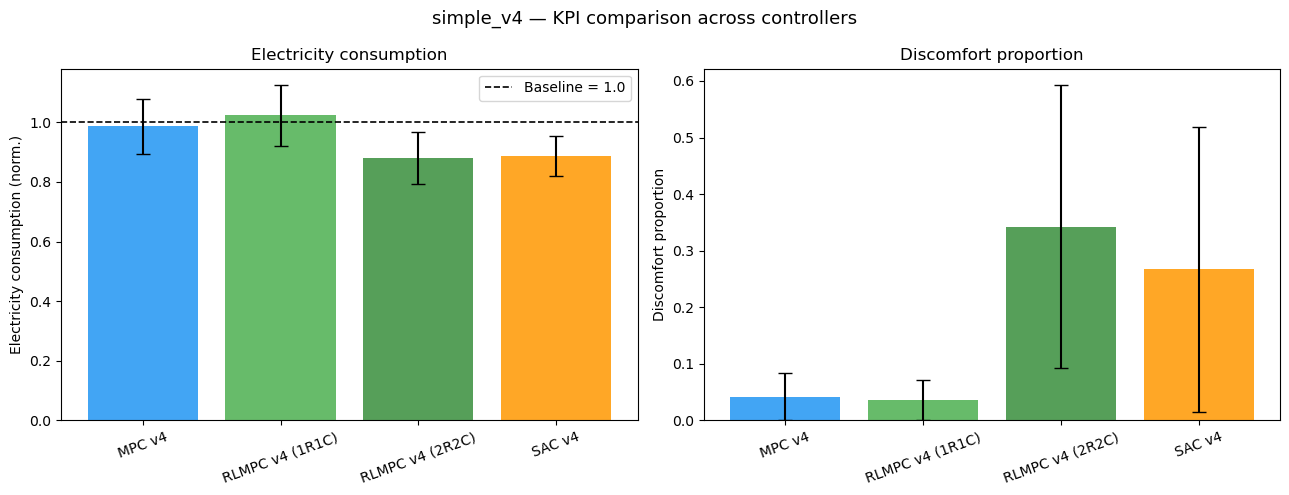

In [3]:
# ── Bar chart comparison ─────────────────────────────────────────
controllers = ['MPC v4', 'RLMPC v4 (1R1C)', 'RLMPC v4 (2R2C)', 'SAC v4']
dfs = [df_mpc, df_rlmpc, df_2r2c, df_sac]
colors = ['#2196F3', '#4CAF50', '#388E3C', '#FF9800']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# electricity
elec_means = [df['electricity_consumption_total'].mean() if not df.empty else float('nan') for df in dfs]
elec_stds  = [df['electricity_consumption_total'].std()  if not df.empty else 0.0 for df in dfs]
axes[0].bar(controllers, elec_means, yerr=elec_stds, color=colors, capsize=5, alpha=0.85)
axes[0].axhline(1.0, color='black', ls='--', lw=1.2, label='Baseline = 1.0')
axes[0].set_ylabel('Electricity consumption (norm.)'); axes[0].set_title('Electricity consumption')
axes[0].legend(); axes[0].tick_params(axis='x', rotation=20)

# discomfort
disc_means = [df['discomfort_proportion'].mean() if not df.empty else float('nan') for df in dfs]
disc_stds  = [df['discomfort_proportion'].std()  if not df.empty else 0.0 for df in dfs]
axes[1].bar(controllers, disc_means, yerr=disc_stds, color=colors, capsize=5, alpha=0.85)
axes[1].set_ylabel('Discomfort proportion'); axes[1].set_title('Discomfort proportion')
axes[1].tick_params(axis='x', rotation=20)

fig.suptitle('simple_v4 — KPI comparison across controllers', fontsize=13)
fig.tight_layout()

fdir = REPO / 'figures' / 'simple_v4_comparison'
fdir.mkdir(parents=True, exist_ok=True)
fig.savefig(fdir / 'kpi_bar_comparison.png', dpi=120, bbox_inches='tight')
plt.show()


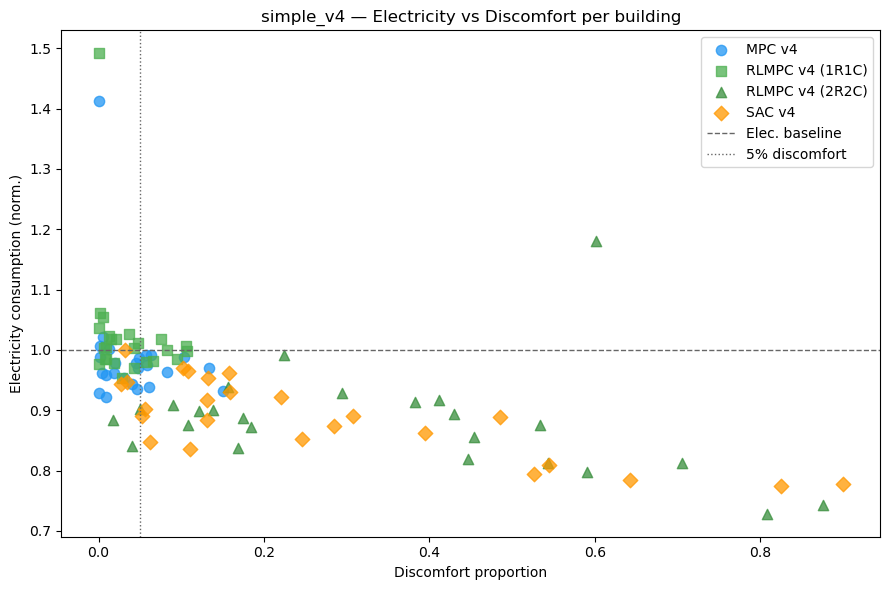

In [4]:
# ── Per-building scatter: electricity vs discomfort ──────────────
fig, ax = plt.subplots(figsize=(9, 6))
markers = ['o', 's', '^', 'D']
for (name, df, c, m) in zip(controllers, dfs, colors, markers):
    if df.empty:
        continue
    ax.scatter(df['discomfort_proportion'], df['electricity_consumption_total'],
               color=c, marker=m, s=55, alpha=0.75, label=name)

ax.axhline(1.0, color='0.4', ls='--', lw=1, label='Elec. baseline')
ax.axvline(0.05, color='0.4', ls=':', lw=1, label='5% discomfort')
ax.set_xlabel('Discomfort proportion'); ax.set_ylabel('Electricity consumption (norm.)')
ax.set_title('simple_v4 — Electricity vs Discomfort per building')
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig(fdir / 'elec_vs_discomfort_scatter.png', dpi=120, bbox_inches='tight')
plt.show()


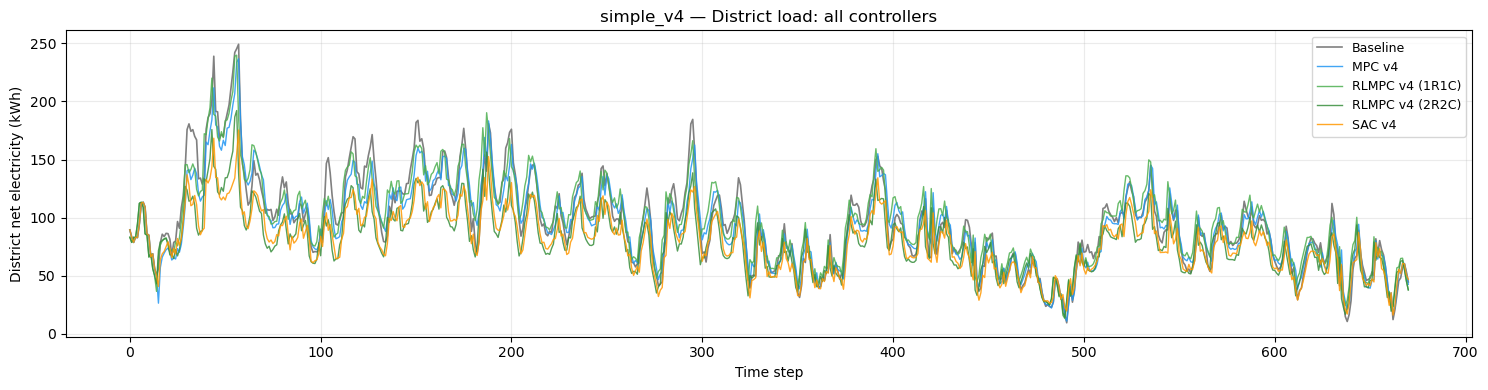

In [5]:
# ── District load comparison: all controllers ────────────────────
from src.district_analysis import aggregate_controller_rollouts, load_or_run_citylearn_baseline_district

BL_DIR = RESULTS / 'raw' / 'citylearn_baseline' / 'no_occupant' / 'baseline'
BL_SUM = RESULTS / 'summaries' / 'citylearn_baseline' / 'no_occupant'
baseline_district = load_or_run_citylearn_baseline_district(output_dir=BL_DIR, summary_dir=BL_SUM)

ctrl_configs = [
    ('MPC v4',           'mpc',        'simple_v4'),
    ('RLMPC v4 (1R1C)',  'rlmpc',      'simple_v4_1r1c'),
    ('RLMPC v4 (2R2C)',  'rlmpc',      'simple_v4'),
    ('SAC v4',           'sac_merlin', 'baseline'),
]

n = len(baseline_district)
compare_load = pd.DataFrame({'time_step': np.arange(n),
                              'Baseline': baseline_district['net_electricity_consumption'].values})

for label, ctrl, case in ctrl_configs:
    d, missing = aggregate_controller_rollouts(
        controller=ctrl, case=case, results_root=RESULTS, buildings=BUILDINGS)
    if not missing and len(d) > 0:
        compare_load[label] = d['net_electricity_consumption'].iloc[:n].values
    else:
        print(f"  {label}: {len(missing)} missing rollouts")

fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(compare_load['time_step'], compare_load['Baseline'], color='0.5', lw=1.2, label='Baseline')
for label, color in zip([x[0] for x in ctrl_configs], colors):
    if label in compare_load.columns:
        ax.plot(compare_load['time_step'], compare_load[label], color=color, lw=1.0, alpha=0.85, label=label)
ax.set_xlabel('Time step'); ax.set_ylabel('District net electricity (kWh)')
ax.legend(fontsize=9)
ax.grid(alpha=0.25); ax.set_title('simple_v4 — District load: all controllers')
fig.tight_layout()
fig.savefig(fdir / 'district_load_timeseries_multi.png', dpi=120, bbox_inches='tight')
plt.show()


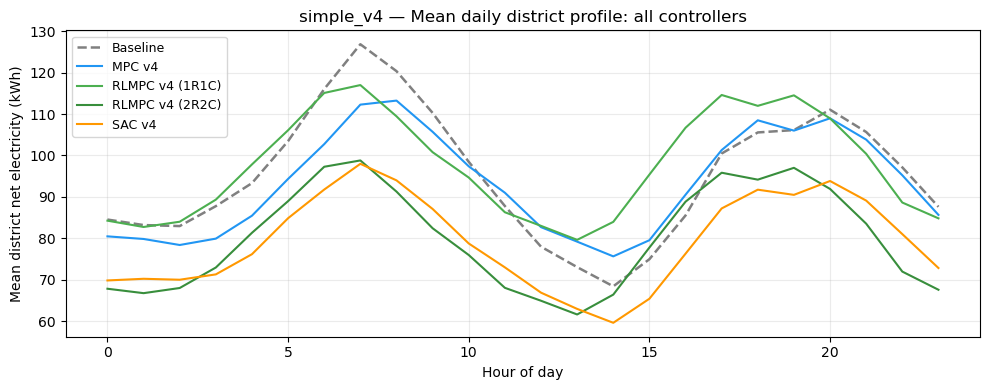

In [6]:
# ── Mean daily district profile comparison ───────────────────────
feb_steps = 672
n2 = min(feb_steps, len(compare_load))
hours = np.arange(n2) % 24

fig, ax = plt.subplots(figsize=(10, 4))
bl_mean = compare_load['Baseline'].iloc[:n2].groupby(hours).mean()
ax.plot(bl_mean.index, bl_mean.values, color='0.5', lw=1.8, ls='--', label='Baseline')

for label, color in zip([x[0] for x in ctrl_configs], colors):
    if label in compare_load.columns:
        col_mean = compare_load[label].iloc[:n2].groupby(hours).mean()
        ax.plot(col_mean.index, col_mean.values, color=color, lw=1.5, label=label)

ax.set_xlabel('Hour of day'); ax.set_ylabel('Mean district net electricity (kWh)')
ax.legend(fontsize=9)
ax.grid(alpha=0.25); ax.set_title('simple_v4 — Mean daily district profile: all controllers')
fig.tight_layout()
fig.savefig(fdir / 'district_mean_daily_profile_multi.png', dpi=120, bbox_inches='tight')
plt.show()


In [7]:
# ── Summary table with all KPIs side by side ─────────────────────
summary_rows = []
for name, df in zip(controllers, dfs):
    if df.empty:
        continue
    summary_rows.append({
        'Controller': name,
        'n_buildings': len(df),
        'elec_mean':   df['electricity_consumption_total'].mean(),
        'elec_median': df['electricity_consumption_total'].median(),
        'disc_mean':   df['discomfort_proportion'].mean(),
        'disc_median': df['discomfort_proportion'].median(),
        'disc_cold_mean': df['discomfort_cold_proportion'].mean(),
        'disc_hot_mean':  df['discomfort_hot_proportion'].mean() if 'discomfort_hot_proportion' in df else float('nan'),
        'peak_mean':   df['daily_peak_average'].mean(),
    })

summary = pd.DataFrame(summary_rows).set_index('Controller')
display(Markdown('### Full KPI summary'))
display(summary.round(4))


### Full KPI summary

,n_buildings,elec_mean,elec_median,disc_mean,disc_median,disc_cold_mean,disc_hot_mean,peak_mean
Controller,,,,,,,,
MPC v4,25,0.9864,0.9707,0.0420,0.0399,0.0387,0.0033,1.0160
RLMPC v4 (1R1C),25,1.0230,1.0035,0.0358,0.0213,0.0238,0.0120,1.0346
RLMPC v4 (2R2C),25,0.8806,0.8838,0.3421,0.2947,0.3164,0.0258,0.9677
SAC v4,25,0.8870,0.8900,0.2668,0.1573,0.2529,0.0139,0.9652


---
## SAC v4 fixed — `simple_v4_ramp01`

Two bugs fixed versus the original SAC v4 run:
1. **Setpoint bias removed** — reward now tracks $T^{sp}$ directly (`tsp_lower_bias=0.0`), not $T^{sp}-0.5$.
2. **Action smoothness penalty added** — ramp term $0.1 \cdot (u_k - u_{k-1})^2$ suppresses bang-bang heating.

Updated cost signal per building:

$$J_k = \frac{1.5 \cdot (T_k - T^{sp}_k)^2}{(2\,°C)^2} + 1.0 \cdot \lambda_k \cdot u_k + 0.1 \cdot (u_k - u_{k-1})^2$$

| Controller | Case label | tsp\_bias | ramp\_weight |
|---|---|---|---|
| **SAC v4 (old)** | `simple_v4` | 0.5 | 0.0 |
| **SAC v4 fixed** | `simple_v4_ramp01` | 0.0 | 0.1 |

In [ ]:
def load_sac_case(case_label):
    rows = []
    for f in sorted(glob.glob(str(RESULTS / 'summaries/sac_merlin/building_*/no_occupant/summary.csv'))):
        try:
            df = pd.read_csv(f)
            if 'case' in df.columns:
                sub = df[df['case'] == case_label]
                if len(sub):
                    rows.append(sub)
        except Exception:
            pass
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

df_sac_old   = load_sac_case('simple_v4')     # old: tsp_bias=0.5, no ramp
df_sac_fixed = load_sac_case('simple_v4_ramp01')  # fixed: tsp_bias=0.0, ramp=0.1

print(f"SAC v4 (old):   {len(df_sac_old)} buildings")
print(f"SAC v4 fixed:   {len(df_sac_fixed)} buildings")
if not df_sac_fixed.empty and 'simple_v4_tsp_lower_bias' in df_sac_fixed.columns:
    print(f"  tsp_lower_bias = {df_sac_fixed['simple_v4_tsp_lower_bias'].iloc[0]}")
if not df_sac_fixed.empty and 'simple_v4_ramp_weight' in df_sac_fixed.columns:
    print(f"  ramp_weight    = {df_sac_fixed['simple_v4_ramp_weight'].iloc[0]}")

In [ ]:
# ── KPI table: fixed vs old SAC + reference controllers ──────────
controllers_r = ['MPC v4', 'RLMPC v4 (1R1C)', 'SAC v4 (old)', 'SAC v4 fixed']
dfs_r         = [df_mpc,   df_rlmpc,           df_sac_old,     df_sac_fixed]
colors_r      = ['#2196F3', '#4CAF50',           '#FF9800',       '#E53935']

summary_rows = []
for name, df in zip(controllers_r, dfs_r):
    if df.empty:
        summary_rows.append({'Controller': name, 'n_buildings': 0,
                              'elec_mean': float('nan'), 'elec_median': float('nan'),
                              'disc_mean': float('nan'), 'disc_median': float('nan'),
                              'disc_cold_mean': float('nan'), 'disc_hot_mean': float('nan'),
                              'peak_mean': float('nan')})
        continue
    summary_rows.append({
        'Controller':    name,
        'n_buildings':   len(df),
        'elec_mean':     df['electricity_consumption_total'].mean(),
        'elec_median':   df['electricity_consumption_total'].median(),
        'disc_mean':     df['discomfort_proportion'].mean(),
        'disc_median':   df['discomfort_proportion'].median(),
        'disc_cold_mean': df['discomfort_cold_proportion'].mean(),
        'disc_hot_mean': df['discomfort_hot_proportion'].mean() if 'discomfort_hot_proportion' in df else float('nan'),
        'peak_mean':     df['daily_peak_average'].mean(),
    })

summary_r = pd.DataFrame(summary_rows).set_index('Controller')
display(Markdown('### KPI summary — SAC v4 fixed vs reference controllers'))
display(summary_r.round(4))

In [ ]:
# ── Bar chart: fixed SAC vs reference ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

elec_means = [df['electricity_consumption_total'].mean() if not df.empty else float('nan') for df in dfs_r]
elec_stds  = [df['electricity_consumption_total'].std()  if not df.empty else 0.0 for df in dfs_r]
axes[0].bar(controllers_r, elec_means, yerr=elec_stds, color=colors_r, capsize=5, alpha=0.85)
axes[0].axhline(1.0, color='black', ls='--', lw=1.2, label='Baseline = 1.0')
axes[0].set_ylabel('Electricity consumption (norm.)'); axes[0].set_title('Electricity consumption')
axes[0].legend(); axes[0].tick_params(axis='x', rotation=20)

disc_means = [df['discomfort_proportion'].mean() if not df.empty else float('nan') for df in dfs_r]
disc_stds  = [df['discomfort_proportion'].std()  if not df.empty else 0.0 for df in dfs_r]
axes[1].bar(controllers_r, disc_means, yerr=disc_stds, color=colors_r, capsize=5, alpha=0.85)
axes[1].set_ylabel('Discomfort proportion'); axes[1].set_title('Discomfort proportion')
axes[1].tick_params(axis='x', rotation=20)

fig.suptitle('simple_v4 fixed — KPI comparison', fontsize=13)
fig.tight_layout()

fdir_r = REPO / 'figures' / 'simple_v4_ramp01'
fdir_r.mkdir(parents=True, exist_ok=True)
fig.savefig(fdir_r / 'kpi_bar_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Per-building scatter ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 6))
markers_r = ['o', 's', 'D', '*']
for (name, df, c, m) in zip(controllers_r, dfs_r, colors_r, markers_r):
    if df.empty:
        continue
    ax.scatter(df['discomfort_proportion'], df['electricity_consumption_total'],
               color=c, marker=m, s=60 if m != '*' else 90, alpha=0.75, label=name)

ax.axhline(1.0, color='0.4', ls='--', lw=1, label='Elec. baseline')
ax.axvline(0.05, color='0.4', ls=':', lw=1, label='5% discomfort')
ax.set_xlabel('Discomfort proportion'); ax.set_ylabel('Electricity consumption (norm.)')
ax.set_title('simple_v4 fixed — Electricity vs Discomfort per building')
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig(fdir_r / 'elec_vs_discomfort_scatter.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
# ── District load + mean daily profile: fixed SAC vs reference ───
from src.district_analysis import aggregate_controller_rollouts, load_or_run_citylearn_baseline_district

ctrl_configs_r = [
    ('MPC v4',           'mpc',        'simple_v4'),
    ('RLMPC v4 (1R1C)',  'rlmpc',      'simple_v4_1r1c'),
    ('SAC v4 (old)',     'sac_merlin', 'simple_v4'),
    ('SAC v4 fixed',     'sac_merlin', 'simple_v4_ramp01'),
]

baseline_district = load_or_run_citylearn_baseline_district(
    output_dir=RESULTS / 'raw' / 'citylearn_baseline' / 'no_occupant' / 'baseline',
    summary_dir=RESULTS / 'summaries' / 'citylearn_baseline' / 'no_occupant')

n = len(baseline_district)
compare_load_r = pd.DataFrame({'time_step': np.arange(n),
                                'Baseline': baseline_district['net_electricity_consumption'].values})

for lbl, ctrl, case in ctrl_configs_r:
    d, missing = aggregate_controller_rollouts(
        controller=ctrl, case=case, results_root=RESULTS, buildings=BUILDINGS)
    if not missing and len(d) > 0:
        compare_load_r[lbl] = d['net_electricity_consumption'].iloc[:n].values
    else:
        print(f"  {lbl}: {len(missing)} missing rollouts")

# timeseries
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(compare_load_r['time_step'], compare_load_r['Baseline'], color='0.5', lw=1.2, label='Baseline')
for (lbl, _, _), color in zip(ctrl_configs_r, colors_r):
    if lbl in compare_load_r.columns:
        ax.plot(compare_load_r['time_step'], compare_load_r[lbl], color=color, lw=1.0, alpha=0.85, label=lbl)
ax.set_xlabel('Time step'); ax.set_ylabel('District net electricity (kWh)')
ax.legend(fontsize=9); ax.grid(alpha=0.25)
ax.set_title('simple_v4 fixed — District load: all controllers')
fig.tight_layout()
fig.savefig(fdir_r / 'district_load_timeseries_multi.png', dpi=120, bbox_inches='tight')
plt.show()

# mean daily profile
feb_steps = 672
n2 = min(feb_steps, len(compare_load_r))
hours = np.arange(n2) % 24

fig, ax = plt.subplots(figsize=(10, 4))
bl_mean = compare_load_r['Baseline'].iloc[:n2].groupby(hours).mean()
ax.plot(bl_mean.index, bl_mean.values, color='0.5', lw=1.8, ls='--', label='Baseline')
for (lbl, _, _), color in zip(ctrl_configs_r, colors_r):
    if lbl in compare_load_r.columns:
        col_mean = compare_load_r[lbl].iloc[:n2].groupby(hours).mean()
        ax.plot(col_mean.index, col_mean.values, color=color, lw=1.5, label=lbl)
ax.set_xlabel('Hour of day'); ax.set_ylabel('Mean district net electricity (kWh)')
ax.legend(fontsize=9); ax.grid(alpha=0.25)
ax.set_title('simple_v4 fixed — Mean daily district profile')
fig.tight_layout()
fig.savefig(fdir_r / 'district_mean_daily_profile_multi.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
# ── Per-building comfort plots: SAC v4 fixed ─────────────────────
COMFORT_BAND_V4 = 2.0

def plot_comfort_v4(history, ax=None, title=None):
    ax = ax or plt.subplots(figsize=(12, 4))[1]
    x = history['time_step'] if 'time_step' in history.columns else np.arange(len(history))
    tsp = history['effective_setpoint'].to_numpy(dtype=float)
    tin = history['indoor_temperature'].to_numpy(dtype=float)
    lower = tsp - COMFORT_BAND_V4
    upper = tsp + COMFORT_BAND_V4
    ax.plot(x, tin, label='Indoor temp', linewidth=1.5)
    ax.plot(x, tsp, linestyle='--', label='Setpoint', linewidth=1.2, color='tab:orange')
    ax.fill_between(x, lower, upper, color='gray', alpha=0.18, label='±2°C band')
    ax.plot(x, lower, color='gray', alpha=0.35, linewidth=0.7)
    ax.plot(x, upper, color='gray', alpha=0.35, linewidth=0.7)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel('Time step', fontsize=8)
    ax.set_ylabel('Temp [°C]', fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=6)
    return ax

rollout_paths_fixed = sorted(glob.glob(
    str(RESULTS / 'raw/sac_merlin/building_*/no_occupant/simple_v4_ramp01/rollout.csv')))
print(f"Found {len(rollout_paths_fixed)} rollouts")

ncols = 5
nrows = (len(rollout_paths_fixed) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.2, nrows * 3.0), sharey=False)
axes_flat = axes.ravel()

for i, path in enumerate(rollout_paths_fixed):
    df = pd.read_csv(path)
    bname = Path(path).parts[-4]
    plot_comfort_v4(df, ax=axes_flat[i], title=f'SAC fixed — {bname}')

for j in range(i + 1, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle('SAC v4 fixed (simple_v4_ramp01) — comfort all 25 buildings', fontsize=12, y=1.01)
fig.tight_layout()
fdir_r.mkdir(parents=True, exist_ok=True)
fig.savefig(fdir_r / 'sac_merlin_comfort_all25.png', dpi=110, bbox_inches='tight')
plt.show()

![SAC v4 fixed comfort all buildings](../figures/simple_v4_ramp01/sac_merlin_comfort_all25.png)

---
## SAC v4 sym — `simple_v4_sym`

Fix for overheating seen in `simple_v4_ramp01` (buildings 11, 21, 25 had 40–55% hot discomfort).

**Root cause:** `cold_only=True` clipped the comfort penalty to zero whenever `Tin > Tsp`, giving SAC no incentive to avoid overheating. The MPC `simple_v4` stage cost is symmetric — `(Tin − Tsp)² / band²` — and penalises both sides equally.

$$J_k = \frac{1.5 \cdot (T_k - T^{sp}_k)^2}{(2\,°C)^2} + 1.0 \cdot \lambda_k \cdot u_k + 0.1 \cdot (u_k - u_{k-1})^2$$

| Controller | Case label | tsp\_bias | ramp | cold\_only |
|---|---|---|---|---|
| SAC v4 (old) | `simple_v4` | 0.5 | 0.0 | True |
| SAC v4 ramp01 | `simple_v4_ramp01` | 0.0 | 0.1 | True (overheats) |
| **SAC v4 sym** | `simple_v4_sym` | 0.0 | 0.1 | **False** |

In [ ]:
df_sac_sym = load_sac_case('simple_v4_sym')
print(f"SAC v4 sym: {len(df_sac_sym)} buildings")
if not df_sac_sym.empty:
    for col in ['simple_v4_tsp_lower_bias', 'simple_v4_ramp_weight', 'simple_v4_cold_only']:
        if col in df_sac_sym.columns:
            print(f"  {col} = {df_sac_sym[col].iloc[0]}")

controllers_s = ['MPC v4', 'RLMPC v4 (1R1C)', 'SAC v4 (old)', 'SAC v4 ramp01', 'SAC v4 sym']
dfs_s         = [df_mpc,   df_rlmpc,           df_sac_old,     df_sac_fixed,    df_sac_sym]
colors_s      = ['#2196F3', '#4CAF50',           '#FF9800',       '#E53935',       '#9C27B0']

summary_rows = []
for name, df in zip(controllers_s, dfs_s):
    if df.empty:
        continue
    summary_rows.append({
        'Controller':     name,
        'n':              len(df),
        'elec_mean':      df['electricity_consumption_total'].mean(),
        'elec_median':    df['electricity_consumption_total'].median(),
        'disc_mean':      df['discomfort_proportion'].mean(),
        'disc_cold_mean': df['discomfort_cold_proportion'].mean(),
        'disc_hot_mean':  df['discomfort_hot_proportion'].mean() if 'discomfort_hot_proportion' in df else float('nan'),
        'peak_mean':      df['daily_peak_average'].mean(),
    })
display(Markdown('### KPI summary — sym vs ramp01 vs reference'))
display(pd.DataFrame(summary_rows).set_index('Controller').round(4))

In [ ]:
# ── Bar chart: sym vs ramp01 vs reference ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

elec_means = [df['electricity_consumption_total'].mean() if not df.empty else float('nan') for df in dfs_s]
elec_stds  = [df['electricity_consumption_total'].std()  if not df.empty else 0.0 for df in dfs_s]
axes[0].bar(controllers_s, elec_means, yerr=elec_stds, color=colors_s, capsize=5, alpha=0.85)
axes[0].axhline(1.0, color='black', ls='--', lw=1.2, label='Baseline = 1.0')
axes[0].set_ylabel('Electricity consumption (norm.)'); axes[0].set_title('Electricity consumption')
axes[0].legend(); axes[0].tick_params(axis='x', rotation=25)

disc_means = [df['discomfort_proportion'].mean() if not df.empty else float('nan') for df in dfs_s]
disc_stds  = [df['discomfort_proportion'].std()  if not df.empty else 0.0 for df in dfs_s]
axes[1].bar(controllers_s, disc_means, yerr=disc_stds, color=colors_s, capsize=5, alpha=0.85)
axes[1].set_ylabel('Discomfort proportion'); axes[1].set_title('Discomfort proportion')
axes[1].tick_params(axis='x', rotation=25)

fig.suptitle('simple_v4 sym — KPI comparison', fontsize=13)
fig.tight_layout()

fdir_s = REPO / 'figures' / 'simple_v4_sym'
fdir_s.mkdir(parents=True, exist_ok=True)
fig.savefig(fdir_s / 'kpi_bar_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Per-building scatter ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 6))
markers_s = ['o', 's', 'D', '*', 'P']
for (name, df, c, m) in zip(controllers_s, dfs_s, colors_s, markers_s):
    if df.empty:
        continue
    ax.scatter(df['discomfort_proportion'], df['electricity_consumption_total'],
               color=c, marker=m, s=60 if m not in ('*', 'P') else 90, alpha=0.75, label=name)

ax.axhline(1.0, color='0.4', ls='--', lw=1, label='Elec. baseline')
ax.axvline(0.05, color='0.4', ls=':', lw=1, label='5% discomfort')
ax.set_xlabel('Discomfort proportion'); ax.set_ylabel('Electricity consumption (norm.)')
ax.set_title('simple_v4 sym — Electricity vs Discomfort per building')
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig(fdir_s / 'elec_vs_discomfort_scatter.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
# ── District load + mean daily profile: sym vs reference ─────────
ctrl_configs_s = [
    ('MPC v4',           'mpc',        'simple_v4'),
    ('RLMPC v4 (1R1C)',  'rlmpc',      'simple_v4_1r1c'),
    ('SAC v4 (old)',     'sac_merlin', 'simple_v4'),
    ('SAC v4 ramp01',    'sac_merlin', 'simple_v4_ramp01'),
    ('SAC v4 sym',       'sac_merlin', 'simple_v4_sym'),
]

baseline_district = load_or_run_citylearn_baseline_district(
    output_dir=RESULTS / 'raw' / 'citylearn_baseline' / 'no_occupant' / 'baseline',
    summary_dir=RESULTS / 'summaries' / 'citylearn_baseline' / 'no_occupant')

n = len(baseline_district)
compare_load_s = pd.DataFrame({'time_step': np.arange(n),
                                'Baseline': baseline_district['net_electricity_consumption'].values})

for lbl, ctrl, case in ctrl_configs_s:
    d, missing = aggregate_controller_rollouts(
        controller=ctrl, case=case, results_root=RESULTS, buildings=BUILDINGS)
    if not missing and len(d) > 0:
        compare_load_s[lbl] = d['net_electricity_consumption'].iloc[:n].values
    else:
        print(f"  {lbl}: {len(missing)} missing rollouts")

# timeseries
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(compare_load_s['time_step'], compare_load_s['Baseline'], color='0.5', lw=1.2, label='Baseline')
for (lbl, _, _), color in zip(ctrl_configs_s, colors_s):
    if lbl in compare_load_s.columns:
        ax.plot(compare_load_s['time_step'], compare_load_s[lbl], color=color, lw=1.0, alpha=0.85, label=lbl)
ax.set_xlabel('Time step'); ax.set_ylabel('District net electricity (kWh)')
ax.legend(fontsize=9); ax.grid(alpha=0.25)
ax.set_title('simple_v4 sym — District load: all controllers')
fig.tight_layout()
fig.savefig(fdir_s / 'district_load_timeseries_multi.png', dpi=120, bbox_inches='tight')
plt.show()

# mean daily profile
feb_steps = 672
n2 = min(feb_steps, len(compare_load_s))
hours = np.arange(n2) % 24

fig, ax = plt.subplots(figsize=(10, 4))
bl_mean = compare_load_s['Baseline'].iloc[:n2].groupby(hours).mean()
ax.plot(bl_mean.index, bl_mean.values, color='0.5', lw=1.8, ls='--', label='Baseline')
for (lbl, _, _), color in zip(ctrl_configs_s, colors_s):
    if lbl in compare_load_s.columns:
        col_mean = compare_load_s[lbl].iloc[:n2].groupby(hours).mean()
        ax.plot(col_mean.index, col_mean.values, color=color, lw=1.5, label=lbl)
ax.set_xlabel('Hour of day'); ax.set_ylabel('Mean district net electricity (kWh)')
ax.legend(fontsize=9); ax.grid(alpha=0.25)
ax.set_title('simple_v4 sym — Mean daily district profile')
fig.tight_layout()
fig.savefig(fdir_s / 'district_mean_daily_profile_multi.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
# ── Per-building comfort plots: SAC v4 sym ────────────────────────
rollout_paths_sym = sorted(glob.glob(
    str(RESULTS / 'raw/sac_merlin/building_*/no_occupant/simple_v4_sym/rollout.csv')))
print(f"Found {len(rollout_paths_sym)} rollouts")

ncols = 5
nrows = (len(rollout_paths_sym) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4.2, nrows * 3.0), sharey=False)
axes_flat = axes.ravel()

for i, path in enumerate(rollout_paths_sym):
    df = pd.read_csv(path)
    bname = Path(path).parts[-4]
    plot_comfort_v4(df, ax=axes_flat[i], title=f'SAC sym — {bname}')

for j in range(i + 1, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle('SAC v4 sym (simple_v4_sym) — comfort all 25 buildings', fontsize=12, y=1.01)
fig.tight_layout()
fdir_s.mkdir(parents=True, exist_ok=True)
fig.savefig(fdir_s / 'sac_merlin_comfort_all25.png', dpi=110, bbox_inches='tight')
plt.show()

![SAC v4 sym comfort all buildings](../figures/simple_v4_sym/sac_merlin_comfort_all25.png)

## CE1 Time-Biased Setpoint Guard - MPC, GNU-RL/RLMPC, SAC

Run label: `ce1_time_bias_guard_1c_1r1c`

Cost/reward used for the new GNU-RL/RLMPC and SAC runs:

`J_k = 0.5 * [3*((Tin-(Tsp+bias))/2)^2 + 60*(cold_guard/1.5)^2 + 15*(hot_guard/2)^2] + 0.5*GridStress*P_heat/5`

`reward = -J_k`, `bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and `cold_guard/hot_guard` are measured against the true setpoint with a `Tsp +/- 2 C` guard. Comfort and time-weighted heating weights sum to 1.0.

GNU-RL/RLMPC uses the same fixed matched inner MPC cost, so PPO cost-parameter updates are skipped. The qpth solver emitted `15035` inaccurate-solution warnings during the full RLMPC run; treat that controller as informative but numerically less clean than explicit MPC/SAC.

Mean building KPIs:

| controller                   | electricity_consumption_total | discomfort_% | cold_%  | hot_%  | kelvin_hours | daily_peak_average |
| ---------------------------- | ----------------------------- | ------------ | ------- | ------ | ------------ | ------------------ |
| MPC time-bias guard          | 1.0237                        | 2.2805       | 1.6344  | 0.6461 | 0.9951       | 1.0207             |
| GNU-RL/RLMPC time-bias guard | 1.0026                        | 3.9225       | 2.4572  | 1.4653 | 0.9906       | 1.0206             |
| SAC time-bias guard          | 0.9131                        | 21.2895      | 18.6329 | 2.6566 | 1.7001       | 0.9750             |

District aggregate KPIs:

| controller                   | total_kwh  | total_vs_citylearn | peak_kwh | peak_vs_citylearn | daily_profile_peak_kwh | daily_profile_peak_hour | ramping_abs_kwh | ramping_vs_citylearn | target_rmse_kwh | above_target_kwh |
| ---------------------------- | ---------- | ------------------ | -------- | ----------------- | ---------------------- | ----------------------- | --------------- | -------------------- | --------------- | ---------------- |
| CityLearn baseline           | 63992.6098 | 1.0000             | 249.2450 | 1.0000            | 126.8675               | 7.0000                  | 6624.5286       | 1.0000               | 38.1714         | 19606.5689       |
| MPC time-bias guard          | 65633.9937 | 1.0256             | 231.1234 | 0.9273            | 110.9644               | 7.0000                  | 6326.9842       | 0.9551               | 35.7940         | 20766.5893       |
| GNU-RL/RLMPC time-bias guard | 63933.2087 | 0.9991             | 226.9578 | 0.9106            | 116.4020               | 16.0000                 | 6586.2066       | 0.9942               | 34.5247         | 19209.4663       |
| SAC time-bias guard          | 55726.5909 | 0.8708             | 175.3356 | 0.7035            | 99.3865                | 7.0000                  | 5429.6185       | 0.8196               | 22.1186         | 11348.4543       |

Weighted term diagnostics:

| controller                   | term                 | mean    | max      |
| ---------------------------- | -------------------- | ------- | -------- |
| GNU-RL/RLMPC time-bias guard | guard_cold           | 0.3163  | 232.8944 |
| GNU-RL/RLMPC time-bias guard | guard_hot            | 0.0171  | 61.8336  |
| GNU-RL/RLMPC time-bias guard | guard_violation_%    | 4.0179  | 100.0000 |
| GNU-RL/RLMPC time-bias guard | mae_to_biased_tref_c | 0.8478  | 7.6052   |
| GNU-RL/RLMPC time-bias guard | mae_to_true_tsp_c    | 0.7147  | 7.7426   |
| GNU-RL/RLMPC time-bias guard | stage_cost           | 1.0460  | 247.8357 |
| GNU-RL/RLMPC time-bias guard | time_weighted_heat   | 0.2812  | 3.2811   |
| GNU-RL/RLMPC time-bias guard | tracking_target      | 0.4314  | 21.6899  |
| MPC time-bias guard          | guard_cold           | 0.2209  | 337.9298 |
| MPC time-bias guard          | guard_hot            | 0.0103  | 67.7810  |
| MPC time-bias guard          | guard_violation_%    | 2.3905  | 100.0000 |
| MPC time-bias guard          | mae_to_biased_tref_c | 0.6762  | 8.0344   |
| MPC time-bias guard          | mae_to_true_tsp_c    | 0.6336  | 8.0125   |
| MPC time-bias guard          | stage_cost           | 0.8109  | 362.1363 |
| MPC time-bias guard          | time_weighted_heat   | 0.2933  | 3.3568   |
| MPC time-bias guard          | tracking_target      | 0.2863  | 24.2066  |
| SAC time-bias guard          | guard_cold           | 5.1401  | 927.0874 |
| SAC time-bias guard          | guard_hot            | 0.4515  | 179.7282 |
| SAC time-bias guard          | guard_violation_%    | 21.7765 | 100.0000 |
| SAC time-bias guard          | mae_to_biased_tref_c | 1.5025  | 11.7906  |
| SAC time-bias guard          | mae_to_true_tsp_c    | 1.4022  | 11.7906  |
| SAC time-bias guard          | stage_cost           | 7.2612  | 969.5229 |
| SAC time-bias guard          | time_weighted_heat   | 0.2394  | 1.6574   |
| SAC time-bias guard          | tracking_target      | 1.4302  | 52.1315  |


![District load](../figures/ce1_time_bias_guard_1c_1r1c_multi/district_load_timeseries_multi.png)

![Mean hourly district profile](../figures/ce1_time_bias_guard_1c_1r1c_multi/district_mean_daily_profile_multi.png)

![Weighted stage-cost terms](../figures/ce1_time_bias_guard_1c_1r1c_multi/weighted_terms_by_controller.png)

![Hourly bias response](../figures/ce1_time_bias_guard_1c_1r1c_multi/hourly_bias_response_multi.png)

## CE1 Time-Biased Setpoint Guard - Full-Action SAC Ablation

Run labels: `ce1_time_bias_guard_1c_1r1c` for MPC/GNU-RL/RLMPC/clipped SAC; `ce1_time_bias_guard_1c_1r1c_a1` for full-action SAC; `ce1_time_bias_guard_1c_1r1c_mpcjs15_a1` for SAC with a January MPC jump-start and 15 training episodes; `ce1_time_bias_guard_1c_1r1c_bc_mpc_only_es_a1` for PI + MPC behavior cloning only; `ce1_time_bias_guard_1c_1r1c_bc_mpc_sac10_es_a1` for PI + MPC behavior cloning + 10 SAC reward-training episodes; `ce1_time_bias_guard_1c_1r1c_sac_exp_shield_auto_a1` for PI jump-start + 10 SAC reward-training episodes with structured exploration, learned entropy alpha, and a cold comfort shield.

Cost/reward used for the new GNU-RL/RLMPC and SAC runs:

`J_k = 0.5 * [3*((Tin-(Tsp+bias))/2)^2 + 60*(cold_guard/1.5)^2 + 15*(hot_guard/2)^2] + 0.5*GridStress*P_heat/5`

`reward = -J_k`, `bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and `cold_guard/hot_guard` are measured against the true setpoint with a `Tsp +/- 2 C` guard. Comfort and time-weighted heating weights sum to 1.0.

GNU-RL/RLMPC uses the same fixed matched inner MPC cost, so PPO cost-parameter updates are skipped. The qpth solver emitted `0` inaccurate-solution warnings during the full RLMPC run; treat that controller as informative but numerically less clean than explicit MPC/SAC.

The full-action SAC row uses the same MERLIN-style pipeline and reward as clipped SAC, with only `action_scaling_coefficient=1.0` instead of `0.5`. The MPC jump-start SAC row replaces the first January PI exploration episode with actions generated by the same 1R1C time-bias MPC teacher, then trains SAC for the remaining episodes. The BC rows keep the January PI replay episode, train the SAC actor offline against January MPC action labels with validation early stopping (`patience=5`), then either deploy immediately or continue with 10 SAC reward-training episodes before February deployment. The exploration/shield SAC row removes MPC behavior cloning, learns the entropy coefficient (`target_entropy=-1`), replaces some SAC actions with structured random high-heat exploration during January reward training, and applies a PI-style heating floor when `Tin < Tsp - 2 C` during training and February deployment.

Mean building KPIs:

| controller                                                          | electricity_consumption_total | discomfort_% | cold_%  | hot_%  | kelvin_hours | daily_peak_average |
| ------------------------------------------------------------------- | ----------------------------- | ------------ | ------- | ------ | ------------ | ------------------ |
| GNU-RL/RLMPC time-bias guard                                        | 1.0026                        | 3.9225       | 2.4572  | 1.4653 | 0.9906       | 1.0206             |
| SAC time-bias guard (actor 0-0.5)                                   | 0.9131                        | 21.2895      | 18.6329 | 2.6566 | 1.7001       | 0.9750             |
| SAC time-bias guard (actor 0-1)                                     | 0.9317                        | 19.1427      | 15.5964 | 3.5464 | 1.6589       | 0.9981             |
| SAC time-bias guard (MPC jump-start, 15 ep, actor 0-1)              | 0.9081                        | 21.9015      | 20.5416 | 1.3600 | 1.6807       | 0.9806             |
| SAC BC-only from MPC (PI+BC, actor 0-1)                             | 0.8373                        | 35.8125      | 35.3498 | 0.4626 | 2.7820       | 0.9306             |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1)                    | 0.9332                        | 19.3099      | 15.7220 | 3.5879 | 1.6507       | 0.9975             |
| SAC MERLIN structured exploration + shield + auto-alpha (actor 0-1) | 0.9194                        | 14.1039      | 7.6101  | 6.4938 | 1.4462       | 1.1035             |

District aggregate KPIs:

| controller                                                          | total_kwh  | total_vs_citylearn | peak_kwh | peak_vs_citylearn | daily_profile_peak_kwh | daily_profile_peak_hour | ramping_abs_kwh | ramping_vs_citylearn | target_rmse_kwh | above_target_kwh |
| ------------------------------------------------------------------- | ---------- | ------------------ | -------- | ----------------- | ---------------------- | ----------------------- | --------------- | -------------------- | --------------- | ---------------- |
| CityLearn baseline                                                  | 63992.6098 | 1.0000             | 249.2450 | 1.0000            | 126.8675               | 7.0000                  | 6624.5286       | 1.0000               | 38.1714         | 19606.5689       |
| MPC time-bias guard                                                 | 65633.9937 | 1.0256             | 231.1234 | 0.9273            | 110.9644               | 7.0000                  | 6326.9842       | 0.9551               | 35.7940         | 20766.5893       |
| GNU-RL/RLMPC time-bias guard                                        | 63933.2087 | 0.9991             | 226.9578 | 0.9106            | 116.4020               | 16.0000                 | 6586.2066       | 0.9942               | 34.5247         | 19209.4663       |
| SAC time-bias guard (actor 0-0.5)                                   | 55726.5909 | 0.8708             | 175.3356 | 0.7035            | 99.3865                | 7.0000                  | 5429.6185       | 0.8196               | 22.1186         | 11348.4543       |
| SAC time-bias guard (actor 0-1)                                     | 57824.3388 | 0.9036             | 208.4101 | 0.8362            | 105.2449               | 7.0000                  | 5658.3319       | 0.8541               | 25.6749         | 13350.5711       |
| SAC time-bias guard (MPC jump-start, 15 ep, actor 0-1)              | 55365.9190 | 0.8652             | 192.7407 | 0.7733            | 95.7331                | 7.0000                  | 5460.3075       | 0.8243               | 22.2737         | 11180.8897       |
| SAC BC-only from MPC (PI+BC, actor 0-1)                             | 48875.6479 | 0.7638             | 172.4377 | 0.6918            | 83.8271                | 20.0000                 | 5147.0924       | 0.7770               | 16.2243         | 6171.6569        |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1)                    | 57966.3764 | 0.9058             | 204.0310 | 0.8186            | 107.0352               | 7.0000                  | 5720.6311       | 0.8636               | 26.2167         | 13566.7375       |
| SAC MERLIN structured exploration + shield + auto-alpha (actor 0-1) | 56866.4853 | 0.8886             | 214.0687 | 0.8589            | 112.0478               | 7.0000                  | 8115.3011       | 1.2250               | 27.1916         | 13078.2383       |

Weighted term diagnostics:

| controller                                                          | term                 | mean     | max       |
| ------------------------------------------------------------------- | -------------------- | -------- | --------- |
| GNU-RL/RLMPC time-bias guard                                        | guard_cold           | 0.3163   | 232.8944  |
| GNU-RL/RLMPC time-bias guard                                        | guard_hot            | 0.0171   | 61.8336   |
| GNU-RL/RLMPC time-bias guard                                        | guard_violation_%    | 4.0179   | 100.0000  |
| GNU-RL/RLMPC time-bias guard                                        | mae_to_biased_tref_c | 0.8478   | 7.6052    |
| GNU-RL/RLMPC time-bias guard                                        | mae_to_true_tsp_c    | 0.7147   | 7.7426    |
| GNU-RL/RLMPC time-bias guard                                        | stage_cost           | 1.0460   | 247.8357  |
| GNU-RL/RLMPC time-bias guard                                        | time_weighted_heat   | 0.2812   | 3.2811    |
| GNU-RL/RLMPC time-bias guard                                        | tracking_target      | 0.4314   | 21.6899   |
| MPC time-bias guard                                                 | guard_cold           | 0.2209   | 337.9298  |
| MPC time-bias guard                                                 | guard_hot            | 0.0103   | 67.7810   |
| MPC time-bias guard                                                 | guard_violation_%    | 2.3905   | 100.0000  |
| MPC time-bias guard                                                 | mae_to_biased_tref_c | 0.6762   | 8.0344    |
| MPC time-bias guard                                                 | mae_to_true_tsp_c    | 0.6336   | 8.0125    |
| MPC time-bias guard                                                 | stage_cost           | 0.8109   | 362.1363  |
| MPC time-bias guard                                                 | time_weighted_heat   | 0.2933   | 3.3568    |
| MPC time-bias guard                                                 | tracking_target      | 0.2863   | 24.2066   |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1)                    | guard_cold           | 1.7397   | 598.6582  |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1)                    | guard_hot            | 1.4985   | 665.4878  |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1)                    | guard_violation_%    | 19.8629  | 100.0000  |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1)                    | mae_to_biased_tref_c | 1.4573   | 21.4579   |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1)                    | mae_to_true_tsp_c    | 1.3482   | 20.8395   |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1)                    | stage_cost           | 4.9794   | 829.7375  |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1)                    | time_weighted_heat   | 0.2544   | 2.6707    |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1)                    | tracking_target      | 1.4868   | 172.6659  |
| SAC BC-only from MPC (PI+BC, actor 0-1)                             | guard_cold           | 108.9694 | 4543.7988 |
| SAC BC-only from MPC (PI+BC, actor 0-1)                             | guard_hot            | 0.0025   | 4.5306    |
| SAC BC-only from MPC (PI+BC, actor 0-1)                             | guard_violation_%    | 36.1192  | 100.0000  |
| SAC BC-only from MPC (PI+BC, actor 0-1)                             | mae_to_biased_tref_c | 2.4482   | 19.9770   |
| SAC BC-only from MPC (PI+BC, actor 0-1)                             | mae_to_true_tsp_c    | 2.3870   | 20.4604   |
| SAC BC-only from MPC (PI+BC, actor 0-1)                             | stage_cost           | 114.7793 | 4685.8570 |
| SAC BC-only from MPC (PI+BC, actor 0-1)                             | time_weighted_heat   | 0.1945   | 2.2697    |
| SAC BC-only from MPC (PI+BC, actor 0-1)                             | tracking_target      | 5.6128   | 149.6556  |
| SAC MERLIN structured exploration + shield + auto-alpha (actor 0-1) | guard_cold           | 0.6012   | 369.6581  |
| SAC MERLIN structured exploration + shield + auto-alpha (actor 0-1) | guard_hot            | 1.6183   | 1251.4548 |
| SAC MERLIN structured exploration + shield + auto-alpha (actor 0-1) | guard_violation_%    | 14.0805  | 100.0000  |
| SAC MERLIN structured exploration + shield + auto-alpha (actor 0-1) | mae_to_biased_tref_c | 1.3812   | 26.8349   |
| SAC MERLIN structured exploration + shield + auto-alpha (actor 0-1) | mae_to_true_tsp_c    | 1.2139   | 27.8349   |
| SAC MERLIN structured exploration + shield + auto-alpha (actor 0-1) | stage_cost           | 3.8653   | 1522.4559 |
| SAC MERLIN structured exploration + shield + auto-alpha (actor 0-1) | time_weighted_heat   | 0.2514   | 3.5014    |
| SAC MERLIN structured exploration + shield + auto-alpha (actor 0-1) | tracking_target      | 1.3944   | 270.0421  |
| SAC time-bias guard (MPC jump-start, 15 ep, actor 0-1)              | guard_cold           | 3.0891   | 595.8661  |
| SAC time-bias guard (MPC jump-start, 15 ep, actor 0-1)              | guard_hot            | 0.3944   | 348.5430  |
| SAC time-bias guard (MPC jump-start, 15 ep, actor 0-1)              | guard_violation_%    | 22.0805  | 100.0000  |
| SAC time-bias guard (MPC jump-start, 15 ep, actor 0-1)              | mae_to_biased_tref_c | 1.3817   | 14.6341   |
| SAC time-bias guard (MPC jump-start, 15 ep, actor 0-1)              | mae_to_true_tsp_c    | 1.3361   | 15.6341   |
| SAC time-bias guard (MPC jump-start, 15 ep, actor 0-1)              | stage_cost           | 4.8969   | 631.4998  |
| SAC time-bias guard (MPC jump-start, 15 ep, actor 0-1)              | time_weighted_heat   | 0.2335   | 2.5039    |
| SAC time-bias guard (MPC jump-start, 15 ep, actor 0-1)              | tracking_target      | 1.1799   | 80.3092   |
| SAC time-bias guard (actor 0-0.5)                                   | guard_cold           | 5.1401   | 927.0874  |
| SAC time-bias guard (actor 0-0.5)                                   | guard_hot            | 0.4515   | 179.7282  |
| SAC time-bias guard (actor 0-0.5)                                   | guard_violation_%    | 21.7765  | 100.0000  |
| SAC time-bias guard (actor 0-0.5)                                   | mae_to_biased_tref_c | 1.5025   | 11.7906   |
| SAC time-bias guard (actor 0-0.5)                                   | mae_to_true_tsp_c    | 1.4022   | 11.7906   |
| SAC time-bias guard (actor 0-0.5)                                   | stage_cost           | 7.2612   | 969.5229  |
| SAC time-bias guard (actor 0-0.5)                                   | time_weighted_heat   | 0.2394   | 1.6574    |
| SAC time-bias guard (actor 0-0.5)                                   | tracking_target      | 1.4302   | 52.1315   |
| SAC time-bias guard (actor 0-1)                                     | guard_cold           | 1.4409   | 285.2639  |
| SAC time-bias guard (actor 0-1)                                     | guard_hot            | 1.5783   | 689.4084  |
| SAC time-bias guard (actor 0-1)                                     | guard_violation_%    | 19.5410  | 100.0000  |
| SAC time-bias guard (actor 0-1)                                     | mae_to_biased_tref_c | 1.4422   | 22.0615   |
| SAC time-bias guard (actor 0-1)                                     | mae_to_true_tsp_c    | 1.3408   | 21.1751   |
| SAC time-bias guard (actor 0-1)                                     | stage_cost           | 4.7456   | 865.6373  |
| SAC time-bias guard (actor 0-1)                                     | time_weighted_heat   | 0.2530   | 2.4574    |
| SAC time-bias guard (actor 0-1)                                     | tracking_target      | 1.4735   | 182.5155  |


Behavior-cloning loss summary:

| controller                                       | epoch   | bc_train_loss_mean | bc_train_loss_max | bc_val_loss_mean | bc_val_loss_max | bc_val_mae_mean | bc_val_abs_error_max |
| ------------------------------------------------ | ------- | ------------------ | ----------------- | ---------------- | --------------- | --------------- | -------------------- |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1) | 87.0000 | 0.0004             | 0.0004            | 0.0010           | 0.0010          | 0.0244          | 0.1260               |
| SAC BC-only from MPC (PI+BC, actor 0-1)          | 87.0000 | 0.0004             | 0.0004            | 0.0010           | 0.0010          | 0.0244          | 0.1260               |


SAC reward-training loss summary by final episode:

| controller                                                          | episode | soft_q1_loss_mean | soft_q1_loss_max | soft_q2_loss_mean | soft_q2_loss_max | policy_loss_mean | policy_loss_max | alpha_loss_mean | alpha_loss_max | alpha_mean | alpha_max | log_pi_mean_mean | log_pi_mean_max | q_new_actions_mean_mean | q_new_actions_mean_max | reward_batch_mean_mean | reward_batch_mean_max |
| ------------------------------------------------------------------- | ------- | ----------------- | ---------------- | ----------------- | ---------------- | ---------------- | --------------- | --------------- | -------------- | ---------- | --------- | ---------------- | --------------- | ----------------------- | ---------------------- | ---------------------- | --------------------- |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1)                    | 10.0000 | 0.2261            | 4.1044           | 0.2271            | 3.5264           | -55.4326         | 15.9619         |                 |                |            |           | 0.9399           | 1.6856          | 56.1846                 | 198.7063               | 1.3354                 | 4.3580                |
| SAC MERLIN structured exploration + shield + auto-alpha (actor 0-1) | 10.0000 | 2.4016            | 29.9835          | 2.4121            | 28.5109          | 86.2529          | 1264.2410       | 0.0013          | 0.9915         | 3.1369     | 22.4704   | 0.9980           | 1.4165          | -83.1263                | 203.8437               | -3.2141                | 3.8659                |


Online reward summary:

| controller                        | episode | phase          | reward_mean | reward_sum    | reward_min  |
| --------------------------------- | ------- | -------------- | ----------- | ------------- | ----------- |
| SAC time-bias guard (actor 0-0.5) | 1.0000  | sac_training   | -68.3279    | -1267481.7225 | -4628.1894  |
| SAC time-bias guard (actor 0-0.5) | 2.0000  | sac_training   | -21.5449    | -400196.4480  | -6835.9819  |
| SAC time-bias guard (actor 0-0.5) | 3.0000  | sac_training   | -16.6054    | -308445.7705  | -1559.6303  |
| SAC time-bias guard (actor 0-0.5) | 4.0000  | sac_training   | -16.7988    | -312037.8078  | -1603.9027  |
| SAC time-bias guard (actor 0-0.5) | 5.0000  | sac_training   | -16.1715    | -300385.8422  | -3029.8549  |
| SAC time-bias guard (actor 0-0.5) | 6.0000  | sac_training   | -15.6694    | -291059.7018  | -1272.0418  |
| SAC time-bias guard (actor 0-0.5) | 7.0000  | sac_training   | -15.7957    | -293404.9033  | -1731.8690  |
| SAC time-bias guard (actor 0-0.5) | 8.0000  | sac_training   | -16.0838    | -298755.8205  | -1555.5528  |
| SAC time-bias guard (actor 0-0.5) | 9.0000  | sac_training   | -15.5348    | -288558.7168  | -1560.1686  |
| SAC time-bias guard (actor 0-1)   | 0.0000  | pi_exploration | -110.9276   | -2060480.1769 | -18613.8767 |
| SAC time-bias guard (actor 0-1)   | 1.0000  | pi_exploration | -1.0495     | -26.2369      | -1.8741     |
| SAC time-bias guard (actor 0-1)   | 1.0000  | sac_training   | -49.6363    | -920754.1113  | -4257.0514  |
| SAC time-bias guard (actor 0-1)   | 2.0000  | sac_training   | -13.1697    | -244627.4641  | -1503.2822  |
| SAC time-bias guard (actor 0-1)   | 3.0000  | sac_training   | -11.2065    | -208161.3068  | -940.7583   |
| SAC time-bias guard (actor 0-1)   | 4.0000  | sac_training   | -10.0283    | -186275.6250  | -1291.2842  |
| SAC time-bias guard (actor 0-1)   | 5.0000  | sac_training   | -9.9771     | -185324.1779  | -1250.7244  |
| SAC time-bias guard (actor 0-1)   | 6.0000  | sac_training   | -9.1867     | -170642.2740  | -1154.2373  |
| SAC time-bias guard (actor 0-1)   | 7.0000  | sac_training   | -9.3994     | -174593.3920  | -921.1903   |
| SAC time-bias guard (actor 0-1)   | 8.0000  | sac_training   | -9.0475     | -168057.6843  | -1038.4542  |
| SAC time-bias guard (actor 0-1)   | 9.0000  | sac_training   | -9.5434     | -177268.4466  | -1208.6700  |


SAC exploration/shield diagnostics by final episode:

| controller                                                          | episode | action_mean | action_max | reward_mean | reward_sum    | policy_action_mean | policy_mean_action_mean | policy_log_std_mean | policy_std_mean | exploration_rate_mean | structured_exploration_applied_mean | structured_exploration_applied_max | comfort_shield_applied_mean | comfort_shield_applied_max | tin_before_action_mean | tsp_before_action_mean |
| ------------------------------------------------------------------- | ------- | ----------- | ---------- | ----------- | ------------- | ------------------ | ----------------------- | ------------------- | --------------- | --------------------- | ----------------------------------- | ---------------------------------- | --------------------------- | -------------------------- | ---------------------- | ---------------------- |
| SAC BC+reward from MPC (PI+BC+10 SAC, actor 0-1)                    | 10.0000 | 0.3177      | 0.9903     | -9.5105     | -176658.0703  |                    |                         |                     |                 |                       | nan                                 | nan                                | nan                         | nan                        |                        |                        |
| SAC BC-only from MPC (PI+BC, actor 0-1)                             | 0.0000  | 0.2113      | 1.0000     | -110.9276   | -2060480.1769 |                    |                         |                     |                 |                       | nan                                 | nan                                | nan                         | nan                        |                        |                        |
| SAC MERLIN structured exploration + shield + auto-alpha (actor 0-1) | 10.0000 | 0.3182      | 1.0000     | -14.6242    | -271645.2669  | 0.2944             | 0.2815                  | -0.9601             | 0.4006          | 0.0500                | 0.04732166890982503                 | True                               | 0.028748317631224766        | True                       | 21.1777                | 19.6817                |
| SAC time-bias guard (MPC jump-start, 15 ep, actor 0-1)              | 14.0000 | 0.3061      | 0.9986     | -0.8697     | -16154.6009   |                    |                         |                     |                 |                       | nan                                 | nan                                | nan                         | nan                        |                        |                        |
| SAC time-bias guard (actor 0-0.5)                                   | 9.0000  | 0.2683      | 0.5000     | -15.5348    | -288558.7168  |                    |                         |                     |                 |                       | nan                                 | nan                                | nan                         | nan                        |                        |                        |
| SAC time-bias guard (actor 0-1)                                     | 9.0000  | 0.3134      | 0.9942     | -9.5434     | -177268.4466  |                    |                         |                     |                 |                       | nan                                 | nan                                | nan                         | nan                        |                        |                        |


![District load](../figures/ce1_time_bias_guard_1c_1r1c_multi/district_load_timeseries_multi.png)

![Mean hourly district profile](../figures/ce1_time_bias_guard_1c_1r1c_multi/district_mean_daily_profile_multi.png)

![Weighted stage-cost terms](../figures/ce1_time_bias_guard_1c_1r1c_multi/weighted_terms_by_controller.png)

![Hourly bias response](../figures/ce1_time_bias_guard_1c_1r1c_multi/hourly_bias_response_multi.png)

![Training diagnostic](../figures/ce1_time_bias_guard_1c_1r1c_multi/bc_training_losses_multi.png)

![Training diagnostic](../figures/ce1_time_bias_guard_1c_1r1c_multi/sac_training_losses_multi.png)

![Training diagnostic](../figures/ce1_time_bias_guard_1c_1r1c_multi/online_training_rewards_multi.png)

![Training diagnostic](../figures/ce1_time_bias_guard_1c_1r1c_multi/sac_exploration_diagnostics_multi.png)

![Reward landscape](../figures/reward_landscape/time_bias_guard_immediate_reward_surface.png)

![Reward landscape](../figures/reward_landscape/time_bias_guard_one_step_proxy_reward_surface_b8_1r1c.png)

![Reward landscape](../figures/reward_landscape/time_bias_guard_reward_vs_action_curves.png)

![Bad-building mean hourly load](../figures/ce1_time_bias_guard_1c_1r1c_idrobust_bad_buildings/bad_building_mean_hourly_load.png)

![Bad-building hourly response](../figures/ce1_time_bias_guard_1c_1r1c_idrobust_bad_buildings/bad_building_hourly_response.png)

![Bad-building weighted terms](../figures/ce1_time_bias_guard_1c_1r1c_idrobust_bad_buildings/bad_building_weighted_terms.png)

<!-- END_BAD_BUILDING_IDROBUST_RC_SECTION -->

## Jan+Feb PI 1R1C Fit - March Holdout

Bad-fitted buildings: `5,8,11,14,19`. PI controlled both fitting months, using Jan+Feb (`0-1415`) for fitting and March (`1416-2159`) as a held-out PI rollout.

The new model is `Jan+Feb PI robust RC`: bounded robust 1R1C fitted on PI-controlled Jan+Feb only. The comparison keeps the former January PI RC and the richer January-ID robust RC.

March holdout fit metrics:

| building    | model                 | one_step_rmse_c | one_step_mae_c | one_step_bias_c | free_run_rmse_c | free_run_mae_c | free_run_bias_c |
| ----------- | --------------------- | --------------- | -------------- | --------------- | --------------- | -------------- | --------------- |
| Building 5  | Former Jan PI RC      | 2.3170          | 1.9896         | -1.5742         | 5.0153          | 4.2379         | -3.8098         |
| Building 5  | Rich Jan ID robust RC | 2.9545          | 2.7111         | -2.6977         | 8.5930          | 8.0983         | -8.0983         |
| Building 5  | Jan+Feb PI robust RC  | 2.0572          | 1.7901         | -0.8766         | 4.0470          | 3.1535         | -2.4300         |
| Building 8  | Former Jan PI RC      | 6.8168          | 4.5470         | 3.9863          | 12.4899         | 11.2340        | 10.9498         |
| Building 8  | Rich Jan ID robust RC | 7.5159          | 4.8597         | 3.9535          | 12.7678         | 10.9729        | 10.6216         |
| Building 8  | Jan+Feb PI robust RC  | 7.7641          | 5.0226         | 4.4437          | 12.7270         | 10.9622        | 10.6868         |
| Building 11 | Former Jan PI RC      | 12.2582         | 11.4454        | -11.0780        | 67.7821         | 63.6841        | -63.6699        |
| Building 11 | Rich Jan ID robust RC | 10.1156         | 9.4759         | -9.1453         | 48.6937         | 45.6521        | -45.6398        |
| Building 11 | Jan+Feb PI robust RC  | 10.3600         | 9.6664         | -9.3870         | 35.1828         | 32.8551        | -32.8123        |
| Building 14 | Former Jan PI RC      | 6.3347          | 5.0981         | 0.8329          | 6.1419          | 5.0576         | 0.9089          |
| Building 14 | Rich Jan ID robust RC | 6.2769          | 4.8678         | 0.3156          | 6.0025          | 4.7762         | 0.3569          |
| Building 14 | Jan+Feb PI robust RC  | 6.2587          | 4.8435         | 0.5803          | 5.9075          | 4.7519         | 0.6906          |
| Building 19 | Former Jan PI RC      | 4.1405          | 3.2592         | 0.1208          | 6.6809          | 5.2410         | 0.4275          |
| Building 19 | Rich Jan ID robust RC | 3.8219          | 2.8966         | 0.3285          | 8.5328          | 6.6386         | 1.6127          |
| Building 19 | Jan+Feb PI robust RC  | 3.8965          | 2.8574         | 0.7950          | 8.3656          | 6.5576         | 3.4037          |

Jan+Feb robust RC training-vs-holdout metrics:

| building    | dataset          | one_step_rmse_c | one_step_bias_c | free_run_rmse_c | free_run_bias_c |
| ----------- | ---------------- | --------------- | --------------- | --------------- | --------------- |
| Building 5  | Jan+Feb PI train | 2.7034          | 0.0025          | 5.7744          | 0.0189          |
| Building 5  | March PI holdout | 2.0572          | -0.8766         | 4.0470          | -2.4300         |
| Building 8  | Jan+Feb PI train | 3.9541          | 0.3841          | 8.1119          | 0.9213          |
| Building 8  | March PI holdout | 7.7641          | 4.4437          | 12.7270         | 10.6868         |
| Building 11 | Jan+Feb PI train | 4.1533          | 0.5325          | 6.4365          | 1.8687          |
| Building 11 | March PI holdout | 10.3600         | -9.3870         | 35.1828         | -32.8123        |
| Building 14 | Jan+Feb PI train | 9.2318          | 0.2880          | 8.5798          | 0.3417          |
| Building 14 | March PI holdout | 6.2587          | 0.5803          | 5.9075          | 0.6906          |
| Building 19 | Jan+Feb PI train | 3.9297          | 0.6670          | 7.2787          | 2.7951          |
| Building 19 | March PI holdout | 3.8965          | 0.7950          | 8.3656          | 3.4037          |

Observed March PI rollout KPIs:

| building    | pi_action_mean | net_electricity_total_kwh | heating_electricity_total_kwh | mae_to_tsp_c | comfort_guard_violation_% | tin_min_c | tin_max_c |
| ----------- | -------------- | ------------------------- | ----------------------------- | ------------ | ------------------------- | --------- | --------- |
| Building 5  | 0.2324         | 3359.0608                 | 2870.3278                     | 3.5810       | 64.8721                   | 14.9026   | 31.8056   |
| Building 8  | 0.1978         | 2762.1256                 | 2143.8647                     | 4.0827       | 61.9112                   | 11.1132   | 42.6020   |
| Building 11 | 0.2124         | 2309.9608                 | 1719.7392                     | 1.8468       | 39.1655                   | 9.5919    | 30.4781   |
| Building 14 | 0.2262         | 1567.1153                 | 1272.6781                     | 7.0404       | 74.5626                   | 5.8371    | 36.4843   |
| Building 19 | 0.2073         | 2418.2004                 | 1803.7449                     | 3.3239       | 58.2773                   | 9.4181    | 40.6220   |


![March one-step RMSE](../figures/jan_feb_pi_robust_march_holdout/march_one_step_rmse.png)

![March free-run RMSE](../figures/jan_feb_pi_robust_march_holdout/march_free_run_rmse.png)

![Training vs holdout](../figures/jan_feb_pi_robust_march_holdout/jan_feb_training_vs_march_holdout.png)

![March PI KPIs](../figures/jan_feb_pi_robust_march_holdout/march_pi_kpis.png)

![Hourly residuals](../figures/jan_feb_pi_robust_march_holdout/march_hourly_residuals.png)

<!-- END_JANFEB_RC_MARCH_HOLDOUT_SECTION -->

## Building 11 2R2C Check + Clean March MPC Comfort

Correction: the previous RC free-run comfort figures were too noisy and not the requested control diagnostic. I removed those image cells from the notebooks. This section uses clean `plot_comfort`-style plots from the actual March MPC rollouts only.

March MPC run:

`ce1_time_bias_guard_1c_1r1c_janfeb_march` using Jan+Feb PI robust 1R1C on bad buildings `5,8,11,14,19`, simulation window `1416-2159`.

Building 11 2R2C fit check:

| dataset          | model                  | one_step_rmse_c | one_step_mae_c | one_step_bias_c | free_run_rmse_c | free_run_mae_c | free_run_bias_c |
| ---------------- | ---------------------- | --------------- | -------------- | --------------- | --------------- | -------------- | --------------- |
| Jan+Feb PI train | Jan+Feb PI robust 1R1C | 4.1533          | 3.0100         | 0.5325          | 6.4365          | 4.8059         | 1.8687          |
| Jan+Feb PI train | Former Jan 2R2C        | 4.5103          | 3.3334         | 0.4831          | 35.7378         | 27.9272        | 3.8218          |
| Jan+Feb PI train | Jan+Feb PI 2R2C        | 4.5536          | 3.3956         | 0.0018          | 46.0387         | 42.3238        | -41.2749        |
| March PI holdout | Jan+Feb PI robust 1R1C | 10.3600         | 9.6664         | -9.3870         | 35.1828         | 32.8551        | -32.8123        |
| March PI holdout | Former Jan 2R2C        | 8.3609          | 7.8523         | -7.5305         | 389.9445        | 348.9756       | -348.9756       |
| March PI holdout | Jan+Feb PI 2R2C        | 8.9125          | 8.3619         | -8.1228         | 419.5549        | 374.1602       | -374.1602       |

March MPC KPIs:

| building    | electricity_consumption_total | daily_peak_average | ramping_average | discomfort_% | cold_% | hot_%  |
| ----------- | ----------------------------- | ------------------ | --------------- | ------------ | ------ | ------ |
| Building 5  | 1.0161                        | 1.0078             | 1.0913          | 0.0000       | 0.0000 | 0.0000 |
| Building 8  | 0.9984                        | 0.9896             | 0.9031          | 7.3095       | 4.1991 | 3.1104 |
| Building 11 | 0.9331                        | 0.9618             | 1.0136          | 10.2384      | 1.4025 | 8.8359 |
| Building 14 | 1.0380                        | 0.9746             | 0.9676          | 4.4547       | 2.1505 | 2.3041 |
| Building 19 | 1.0440                        | 0.9878             | 0.8577          | 5.4004       | 1.8622 | 3.5382 |


![Building 11 2R2C RMSE](../figures/building11_2r2c_march_mpc_comfort/building11_march_2r2c_free_run_rmse.png)

![Building 5 clean MPC comfort](../figures/building11_2r2c_march_mpc_comfort/plot_comfort_mpc_janfeb_rc_march_building_05.png)

![Building 8 clean MPC comfort](../figures/building11_2r2c_march_mpc_comfort/plot_comfort_mpc_janfeb_rc_march_building_08.png)

![Building 11 clean MPC comfort](../figures/building11_2r2c_march_mpc_comfort/plot_comfort_mpc_janfeb_rc_march_building_11.png)

![Building 14 clean MPC comfort](../figures/building11_2r2c_march_mpc_comfort/plot_comfort_mpc_janfeb_rc_march_building_14.png)

![Building 19 clean MPC comfort](../figures/building11_2r2c_march_mpc_comfort/plot_comfort_mpc_janfeb_rc_march_building_19.png)

<!-- END_BUILDING11_2R2C_MARCH_MPC_COMFORT -->

## Fixed 2R2C + Kalman Bad-Building Check

This appends the fixed two-state RC check after adding a Kalman observer for the hidden thermal mass state. The RC parameters are fitted on Jan+Feb PI data for bad buildings `5,8,11,14,19`; March is the rollout holdout.

Files:

- Fixed 2R2C+Kalman models: `results/models/rc/2r2c_*_jan_feb_pi_kalman.json`
- Forecast comparison: `analysis/1r1c_vs_2r2c_kalman_bad_buildings_comparison.csv`
- March MPC KPI comparison: `analysis/march_mpc_1r1c_vs_2r2c_kalman_bad_building_kpis.csv`

March holdout forecast RMSE:

| building    | model                | one_step_rmse_c | horizon_24h_rmse_c | free_run_rmse_c |
| ----------- | -------------------- | --------------- | ------------------ | --------------- |
| Building 5  | 1R1C Jan+Feb robust  | 2.057           | 3.955              | 4.054           |
| Building 5  | 2R2C fixed propagate | 1.979           | 3.632              | 10.504          |
| Building 5  | 2R2C fixed + Kalman  | 1.513           | 2.776              |                 |
| Building 8  | 1R1C Jan+Feb robust  | 7.764           | 12.121             | 12.719          |
| Building 8  | 2R2C fixed propagate | 7.225           | 11.270             | 15.625          |
| Building 8  | 2R2C fixed + Kalman  | 6.561           | 9.200              |                 |
| Building 11 | 1R1C Jan+Feb robust  | 10.360          | 32.704             | 35.209          |
| Building 11 | 2R2C fixed propagate | 6.757           | 18.029             | 221.959         |
| Building 11 | 2R2C fixed + Kalman  | 2.443           | 10.971             |                 |
| Building 14 | 1R1C Jan+Feb robust  | 6.259           | 5.913              | 5.904           |
| Building 14 | 2R2C fixed propagate | 6.289           | 6.111              | 10.157          |
| Building 14 | 2R2C fixed + Kalman  | 6.741           | 5.827              |                 |
| Building 19 | 1R1C Jan+Feb robust  | 3.897           | 7.878              | 8.360           |
| Building 19 | 2R2C fixed propagate | 3.314           | 5.145              | 5.682           |
| Building 19 | 2R2C fixed + Kalman  | 3.207           | 5.157              |                 |

March MPC KPIs:

| building    | model               | electricity_consumption_total | daily_peak_average | ramping_average | discomfort_% | cold_% | hot_% |
| ----------- | ------------------- | ----------------------------- | ------------------ | --------------- | ------------ | ------ | ----- |
| Building 5  | 1R1C Jan+Feb robust | 1.016                         | 1.008              | 1.091           | 0.000        | 0.000  | 0.000 |
| Building 5  | 2R2C fixed + Kalman | 1.016                         | 1.017              | 1.116           | 0.000        | 0.000  | 0.000 |
| Building 8  | 1R1C Jan+Feb robust | 0.998                         | 0.990              | 0.903           | 7.309        | 4.199  | 3.110 |
| Building 8  | 2R2C fixed + Kalman | 0.999                         | 0.990              | 0.904           | 5.910        | 2.799  | 3.110 |
| Building 11 | 1R1C Jan+Feb robust | 0.933                         | 0.962              | 1.014           | 10.238       | 1.403  | 8.836 |
| Building 11 | 2R2C fixed + Kalman | 0.930                         | 0.974              | 1.058           | 2.244        | 0.140  | 2.104 |
| Building 14 | 1R1C Jan+Feb robust | 1.038                         | 0.975              | 0.968           | 4.455        | 2.151  | 2.304 |
| Building 14 | 2R2C fixed + Kalman | 1.031                         | 0.953              | 0.958           | 0.307        | 0.307  | 0.000 |
| Building 19 | 1R1C Jan+Feb robust | 1.044                         | 0.988              | 0.858           | 5.400        | 1.862  | 3.538 |
| Building 19 | 2R2C fixed + Kalman | 1.044                         | 0.994              | 0.877           | 4.469        | 1.304  | 3.166 |

KPI deltas for `2R2C fixed + Kalman - 1R1C Jan+Feb robust`:

| building    | elec_delta | peak_delta | ramp_delta | discomfort_delta_pp | cold_delta_pp | hot_delta_pp |
| ----------- | ---------- | ---------- | ---------- | ------------------- | ------------- | ------------ |
| Building 5  | -0.000     | 0.009      | 0.025      | 0.000               | 0.000         | 0.000        |
| Building 8  | 0.000      | 0.000      | 0.001      | -1.400              | -1.400        | -0.000       |
| Building 11 | -0.003     | 0.012      | 0.045      | -7.994              | -1.262        | -6.732       |
| Building 14 | -0.007     | -0.022     | -0.010     | -4.147              | -1.843        | -2.304       |
| Building 19 | -0.000     | 0.007      | 0.020      | -0.931              | -0.559        | -0.372       |


![march_holdout_24h_forecast_rmse](../figures/2r2c_kalman_bad_buildings/march_holdout_24h_forecast_rmse.png)

![march_mpc_discomfort_comparison](../figures/2r2c_kalman_bad_buildings/march_mpc_discomfort_comparison.png)

![march_mpc_energy_peak_comparison](../figures/2r2c_kalman_bad_buildings/march_mpc_energy_peak_comparison.png)

![march_bad_building_mean_hourly_load](../figures/2r2c_kalman_bad_buildings/march_bad_building_mean_hourly_load.png)

Clean `plot_comfort`-style March MPC comfort plots for the 2R2C+Kalman controller:

![Building 5 2R2C Kalman comfort](../figures/2r2c_kalman_bad_buildings/plot_comfort_2r2c_kalman_march_building_05.png)

![Building 8 2R2C Kalman comfort](../figures/2r2c_kalman_bad_buildings/plot_comfort_2r2c_kalman_march_building_08.png)

![Building 11 2R2C Kalman comfort](../figures/2r2c_kalman_bad_buildings/plot_comfort_2r2c_kalman_march_building_11.png)

![Building 14 2R2C Kalman comfort](../figures/2r2c_kalman_bad_buildings/plot_comfort_2r2c_kalman_march_building_14.png)

![Building 19 2R2C Kalman comfort](../figures/2r2c_kalman_bad_buildings/plot_comfort_2r2c_kalman_march_building_19.png)

<!-- END_2R2C_KALMAN_BAD_BUILDING_CHECK -->

## CE1 Time-Biased Setpoint Guard 2R2C+Kalman - `ce1_time_bias_guard_1c_2r2c_kalman`

Run labels: `ce1_time_bias_guard_1c_2r2c_kalman` for MPC and GNU-RL/RLMPC with January-only 2R2C RC models and a Kalman latent-mass observer; `ce1_time_bias_guard_1c_2r2c_kalman_bc_mpc_only_es_a1` for PI + behavior cloning from the 2R2C+Kalman MPC teacher; `ce1_time_bias_guard_1c_2r2c_kalman_bc_mpc_sac10_es_a1` for the same BC initialization followed by 10 SAC reward-training episodes. Both SAC runs use `action_scaling_coefficient=1.0`.

Cost/reward used for the new GNU-RL/RLMPC and SAC runs:

`J_k = 0.5 * [3*((Tin-(Tsp+bias))/2)^2 + 60*(cold_guard/1.5)^2 + 15*(hot_guard/2)^2] + 0.5*GridStress*P_heat/5`

`reward = -J_k`, `bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and `cold_guard/hot_guard` are measured against the true setpoint with a `Tsp +/- 2 C` guard. Comfort and time-weighted heating weights sum to 1.0.

GNU-RL/RLMPC uses the 2R2C DiffMPC checkpoint trained on January PI data. Because qpth emitted `24148` inaccurate-solution warnings across offline training and February deployment, this row should be treated as informative but numerically less clean than explicit MPC/SAC.

The BC rows keep the January PI replay episode, train the SAC actor offline against January 2R2C+Kalman MPC action labels with validation early stopping (`patience=5`), then either deploy immediately or continue with 10 SAC reward-training episodes before February deployment.

Mean building KPIs:

| controller                                                   | electricity_consumption_total | discomfort_% | cold_%  | hot_%  | kelvin_hours | daily_peak_average |
| ------------------------------------------------------------ | ----------------------------- | ------------ | ------- | ------ | ------------ | ------------------ |
| MPC time-bias guard 2R2C+Kalman                              | 1.0002                        | 1.1418       | 0.8790  | 0.2628 | 0.9785       | 1.0111             |
| GNU-RL/RLMPC time-bias guard 2R2C+Kalman                     | 0.9515                        | 12.1062      | 11.6710 | 0.4353 | 1.5122       | 1.0004             |
| SAC BC-only from 2R2C+Kalman MPC (PI+BC, actor 0-1)          | 0.8683                        | 30.5336      | 30.1850 | 0.3486 | 2.3407       | 0.9444             |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 0.9302                        | 19.1357      | 15.8596 | 3.2761 | 1.6151       | 1.0024             |

District aggregate KPIs:

| controller                                                   | total_kwh  | total_vs_citylearn | peak_kwh | peak_vs_citylearn | daily_profile_peak_kwh | daily_profile_peak_hour | ramping_abs_kwh | ramping_vs_citylearn | target_rmse_kwh | above_target_kwh |
| ------------------------------------------------------------ | ---------- | ------------------ | -------- | ----------------- | ---------------------- | ----------------------- | --------------- | -------------------- | --------------- | ---------------- |
| CityLearn baseline                                           | 63992.6098 | 1.0000             | 249.2450 | 1.0000            | 126.8675               | 7.0000                  | 6624.5286       | 1.0000               | 38.1714         | 19606.5689       |
| MPC time-bias guard 2R2C+Kalman                              | 63876.9888 | 0.9982             | 228.8769 | 0.9183            | 108.0223               | 7.0000                  | 6420.6115       | 0.9692               | 33.8810         | 19073.5796       |
| GNU-RL/RLMPC time-bias guard 2R2C+Kalman                     | 58936.0639 | 0.9210             | 219.9343 | 0.8824            | 108.4848               | 7.0000                  | 6014.6704       | 0.9079               | 28.5040         | 14612.9023       |
| SAC BC-only from 2R2C+Kalman MPC (PI+BC, actor 0-1)          | 51657.2120 | 0.8072             | 182.4352 | 0.7320            | 85.7512                | 7.0000                  | 5113.1798       | 0.7719               | 17.6668         | 8037.1365        |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 57521.5155 | 0.8989             | 204.2400 | 0.8194            | 104.5941               | 7.0000                  | 5664.8013       | 0.8551               | 25.6099         | 13130.3637       |

Weighted term diagnostics:

| controller                                                   | term                 | mean    | max       |
| ------------------------------------------------------------ | -------------------- | ------- | --------- |
| GNU-RL/RLMPC time-bias guard 2R2C+Kalman                     | guard_cold           | 3.2780  | 712.1901  |
| GNU-RL/RLMPC time-bias guard 2R2C+Kalman                     | guard_hot            | 0.0026  | 9.2098    |
| GNU-RL/RLMPC time-bias guard 2R2C+Kalman                     | guard_violation_%    | 12.1848 | 100.0000  |
| GNU-RL/RLMPC time-bias guard 2R2C+Kalman                     | mae_to_biased_tref_c | 1.2357  | 9.6628    |
| GNU-RL/RLMPC time-bias guard 2R2C+Kalman                     | mae_to_true_tsp_c    | 0.9722  | 9.3085    |
| GNU-RL/RLMPC time-bias guard 2R2C+Kalman                     | stage_cost           | 4.4828  | 745.1787  |
| GNU-RL/RLMPC time-bias guard 2R2C+Kalman                     | time_weighted_heat   | 0.2626  | 3.3270    |
| GNU-RL/RLMPC time-bias guard 2R2C+Kalman                     | tracking_target      | 0.9395  | 35.0138   |
| MPC time-bias guard 2R2C+Kalman                              | guard_cold           | 0.0478  | 86.0593   |
| MPC time-bias guard 2R2C+Kalman                              | guard_hot            | 0.0037  | 33.6342   |
| MPC time-bias guard 2R2C+Kalman                              | guard_violation_%    | 1.2280  | 100.0000  |
| MPC time-bias guard 2R2C+Kalman                              | mae_to_biased_tref_c | 0.5583  | 5.2354    |
| MPC time-bias guard 2R2C+Kalman                              | mae_to_true_tsp_c    | 0.6148  | 6.2354    |
| MPC time-bias guard 2R2C+Kalman                              | stage_cost           | 0.5245  | 94.5614   |
| MPC time-bias guard 2R2C+Kalman                              | time_weighted_heat   | 0.2812  | 3.3097    |
| MPC time-bias guard 2R2C+Kalman                              | tracking_target      | 0.1917  | 10.2784   |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | guard_cold           | 1.7168  | 340.1465  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | guard_hot            | 1.0183  | 593.3201  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | guard_violation_%    | 19.5112 | 100.0000  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | mae_to_biased_tref_c | 1.4256  | 18.7887   |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | mae_to_true_tsp_c    | 1.3136  | 19.7887   |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | stage_cost           | 4.3376  | 726.3094  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | time_weighted_heat   | 0.2513  | 2.7392    |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | tracking_target      | 1.3512  | 132.3805  |
| SAC BC-only from 2R2C+Kalman MPC (PI+BC, actor 0-1)          | guard_cold           | 67.5749 | 4121.5621 |
| SAC BC-only from 2R2C+Kalman MPC (PI+BC, actor 0-1)          | guard_hot            | 0.0026  | 5.5267    |
| SAC BC-only from 2R2C+Kalman MPC (PI+BC, actor 0-1)          | guard_violation_%    | 30.7958 | 100.0000  |
| SAC BC-only from 2R2C+Kalman MPC (PI+BC, actor 0-1)          | mae_to_biased_tref_c | 1.9899  | 19.0758   |
| SAC BC-only from 2R2C+Kalman MPC (PI+BC, actor 0-1)          | mae_to_true_tsp_c    | 1.9415  | 19.5817   |
| SAC BC-only from 2R2C+Kalman MPC (PI+BC, actor 0-1)          | stage_cost           | 71.5621 | 4251.1033 |
| SAC BC-only from 2R2C+Kalman MPC (PI+BC, actor 0-1)          | time_weighted_heat   | 0.2099  | 2.2414    |
| SAC BC-only from 2R2C+Kalman MPC (PI+BC, actor 0-1)          | tracking_target      | 3.7747  | 136.4575  |


Behavior-cloning loss summary:

| controller                                                   | epoch   | bc_train_loss_mean | bc_train_loss_max | bc_val_loss_mean | bc_val_loss_max | bc_val_mae_mean | bc_val_abs_error_max |
| ------------------------------------------------------------ | ------- | ------------------ | ----------------- | ---------------- | --------------- | --------------- | -------------------- |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 96.0000 | 0.0004             | 0.0004            | 0.0018           | 0.0018          | 0.0322          | 0.1749               |
| SAC BC-only from 2R2C+Kalman MPC (PI+BC, actor 0-1)          | 96.0000 | 0.0004             | 0.0004            | 0.0018           | 0.0018          | 0.0322          | 0.1749               |


SAC reward-training loss summary by final episode:

| controller                                                   | episode | soft_q1_loss_mean | soft_q1_loss_max | soft_q2_loss_mean | soft_q2_loss_max | policy_loss_mean | policy_loss_max |
| ------------------------------------------------------------ | ------- | ----------------- | ---------------- | ----------------- | ---------------- | ---------------- | --------------- |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 10.0000 | 0.2185            | 3.5104           | 0.2194            | 2.8259           | -55.7632         | 11.3641         |


Online reward summary:

| controller                                                   | episode | phase          | reward_mean | reward_sum    | reward_min  |
| ------------------------------------------------------------ | ------- | -------------- | ----------- | ------------- | ----------- |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 0.0000  | pi_exploration | -110.9276   | -2060480.1769 | -18613.8767 |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 1.0000  | pi_exploration | -1.0495     | -26.2369      | -1.8741     |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 1.0000  | sac_training   | -62.5277    | -1159889.6120 | -5629.6632  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 2.0000  | sac_training   | -12.7118    | -236120.8046  | -1579.2457  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 3.0000  | sac_training   | -10.6111    | -197101.9722  | -1509.0692  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 4.0000  | sac_training   | -10.4660    | -194406.7058  | -1367.8266  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 5.0000  | sac_training   | -9.4990     | -176443.6110  | -1071.9578  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 6.0000  | sac_training   | -9.7097     | -180357.0926  | -1067.5236  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 7.0000  | sac_training   | -9.7373     | -180870.6715  | -1723.6741  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 8.0000  | sac_training   | -9.4820     | -176127.8166  | -1266.8403  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 9.0000  | sac_training   | -8.8503     | -164394.4067  | -1124.8338  |
| SAC BC+reward from 2R2C+Kalman MPC (PI+BC+10 SAC, actor 0-1) | 10.0000 | sac_training   | -9.6395     | -179054.2752  | -975.6228   |
| SAC BC-only from 2R2C+Kalman MPC (PI+BC, actor 0-1)          | 0.0000  | pi_exploration | -110.9276   | -2060480.1769 | -18613.8767 |


![District load](../figures/ce1_time_bias_guard_1c_2r2c_kalman_multi/district_load_timeseries_multi.png)

![Mean hourly district profile](../figures/ce1_time_bias_guard_1c_2r2c_kalman_multi/district_mean_daily_profile_multi.png)

![Weighted stage-cost terms](../figures/ce1_time_bias_guard_1c_2r2c_kalman_multi/weighted_terms_by_controller.png)

![Hourly bias response](../figures/ce1_time_bias_guard_1c_2r2c_kalman_multi/hourly_bias_response_multi.png)

![Training diagnostic](../figures/ce1_time_bias_guard_1c_2r2c_kalman_multi/bc_training_losses_multi.png)

![Training diagnostic](../figures/ce1_time_bias_guard_1c_2r2c_kalman_multi/sac_training_losses_multi.png)

![Training diagnostic](../figures/ce1_time_bias_guard_1c_2r2c_kalman_multi/online_training_rewards_multi.png)

## CE1 Safe-PI Reset MERLIN SAC - `ce1_time_bias_guard_1c_1r1c_sac_safepi_reset_auto_a1`

Run label: `ce1_time_bias_guard_1c_1r1c_sac_safepi_reset_auto_a1`. SAC-only ablation, no MPC teacher and no behavior cloning.

Pipeline: January episode 0 uses the new safe PI replay-fill controller; the following January episodes use SAC reward training. During **all January training phases** (`safe_pi_exploration`, `safe_pi_bootstrap`, and `sac_training`), runaway LSTM temperatures are reset back near the setpoint and that transition is dropped from replay. February deployment is not reset or shielded, so February KPIs are honest deployment results.

SAC settings: `action_scaling_coefficient=1.0`, automatic entropy tuning, robust replay normalization with observation/reward clipping, structured exploration, and cold comfort shield during training. Reward/cost is unchanged:

`J_k = 0.5 * [3*((Tin-(Tsp+bias))/2)^2 + 60*(cold_guard/1.5)^2 + 15*(hot_guard/2)^2] + 0.5*GridStress*P_heat/5`

`reward = -J_k`, `bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and guards use true `Tsp +/- 2 C`.

Mean building KPIs:

| controller | electricity_consumption_total | discomfort_% | cold_% | hot_% | kelvin_hours | daily_peak_average |
| --- | --- | --- | --- | --- | --- | --- |
| SAC time-bias guard (actor 0-0.5) | 0.9131 | 21.2895 | 18.6329 | 2.6566 | 1.7001 | 0.9750 |
| SAC time-bias guard (actor 0-1) | 0.9317 | 19.1427 | 15.5964 | 3.5464 | 1.6589 | 0.9981 |
| SAC structured exploration + shield + auto-alpha | 0.9194 | 14.1039 | 7.6101 | 6.4938 | 1.4462 | 1.1035 |
| SAC 1R1C RC-rollout obs (actor 0-1) | 0.8834 | 31.4896 | 30.2365 | 1.2531 | 1.9482 | 0.9622 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 1.0318 | 21.1026 | 5.3273 | 15.7753 | 1.5594 | 1.0726 |

District aggregate KPIs:

| controller | total_kwh | total_vs_citylearn | peak_kwh | peak_vs_citylearn | daily_profile_peak_kwh | daily_profile_peak_hour | ramping_abs_kwh | ramping_vs_citylearn | target_rmse_kwh | above_target_kwh |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| CityLearn baseline | 63992.6098 | 1.0000 | 249.2450 | 1.0000 | 126.8675 | 7 | 6624.5286 | 1.0000 | 38.1714 | 19606.5689 |
| SAC time-bias guard (actor 0-0.5) | 55726.5909 | 0.8708 | 175.3356 | 0.7035 | 99.3865 | 7 | 5429.6185 | 0.8196 | 22.1186 | 11348.4543 |
| SAC time-bias guard (actor 0-1) | 57824.3388 | 0.9036 | 208.4101 | 0.8362 | 105.2449 | 7 | 5658.3319 | 0.8541 | 25.6749 | 13350.5711 |
| SAC structured exploration + shield + auto-alpha | 56866.4853 | 0.8886 | 214.0687 | 0.8589 | 112.0478 | 7 | 8115.3011 | 1.2250 | 27.1916 | 13078.2383 |
| SAC 1R1C RC-rollout obs (actor 0-1) | 52536.9838 | 0.8210 | 168.9483 | 0.6778 | 94.7193 | 20 | 5551.4101 | 0.8380 | 19.8367 | 9037.9910 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 67679.0857 | 1.0576 | 205.4513 | 0.8243 | 115.9837 | 17 | 6437.0071 | 0.9717 | 37.9966 | 22670.9529 |

New run per-building diagnostics, worst hot discomfort first:

| building | electricity_consumption_total | discomfort_% | cold_% | hot_% | feb_tin_min | feb_tin_max | jan_ep0_tin_min | jan_ep0_tin_max | jan_ep0_raw_next_tin_min | jan_ep0_raw_next_tin_max | reset_steps | replay_dropped_steps | safe_pi_bootstrap_steps |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Building 8 | 1.4553 | 78.5838 | 3.1088 | 75.4750 | 14.8916 | 48.8125 | 14.9372 | 28.5226 | 3.0760 | 60.6892 | 3968 | 3968 | 12 |
| Building 15 | 1.2248 | 52.8090 | 2.4345 | 50.3745 | 13.8624 | 33.2885 | 13.2302 | 21.5069 | 4.8695 | 36.9233 | 2014 | 2014 | 0 |
| Building 22 | 1.3477 | 53.7262 | 7.7990 | 45.9272 | 8.8717 | 45.7215 | 14.0500 | 25.8460 | 11.0656 | 49.6600 | 3379 | 3379 | 0 |
| Building 20 | 1.0175 | 36.2890 | 1.9704 | 34.3186 | 14.4820 | 37.7180 | 14.9924 | 24.6509 | 9.8976 | 35.2613 | 2787 | 2787 | 0 |
| Building 11 | 0.9999 | 29.0271 | 3.0303 | 25.9968 | 17.8649 | 30.1157 | 16.5283 | 25.4953 | -7.6538 | 32.1173 | 2806 | 2806 | 0 |
| Building 21 | 1.0509 | 26.5993 | 0.6734 | 25.9259 | 16.4260 | 33.4178 | 13.2385 | 25.0463 | 11.8956 | 39.4051 | 1228 | 1228 | 0 |
| Building 5 | 1.1475 | 37.6682 | 13.1540 | 24.5142 | 18.1000 | 39.8106 | 18.0801 | 26.9784 | 9.7952 | 39.1685 | 2157 | 2157 | 0 |
| Building 2 | 1.0478 | 40.8669 | 18.5759 | 22.2910 | 15.9822 | 47.0882 | 15.2501 | 24.4811 | 9.5742 | 49.7939 | 2212 | 2212 | 0 |

January safe-PI replay-fill diagnostics:

| building | jan_ep0_tin_min | jan_ep0_tin_max | jan_ep0_raw_next_tin_min | jan_ep0_raw_next_tin_max | reset_steps | replay_dropped_steps | safe_pi_bootstrap_steps |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Building 1 | 13.2739 | 27.1224 | 11.1950 | 35.1303 | 1652 | 1652 | 0 |
| Building 2 | 15.2501 | 24.4811 | 9.5742 | 49.7939 | 2212 | 2212 | 0 |
| Building 3 | 14.0494 | 22.1548 | 13.5758 | 26.9021 | 893 | 893 | 0 |
| Building 4 | 13.2889 | 24.4846 | 11.3427 | 37.6539 | 1060 | 1060 | 0 |
| Building 5 | 18.0801 | 26.9784 | 9.7952 | 39.1685 | 2157 | 2157 | 0 |
| Building 6 | 15.4193 | 25.1133 | 12.3148 | 27.6299 | 1155 | 1155 | 0 |
| Building 7 | 16.0611 | 25.4565 | 11.8366 | 34.9000 | 1416 | 1416 | 0 |
| Building 8 | 14.9372 | 28.5226 | 3.0760 | 60.6892 | 3968 | 3968 | 12 |
| Building 9 | 13.3614 | 28.3414 | 10.7855 | 37.7597 | 755 | 755 | 0 |
| Building 10 | 13.3163 | 22.2110 | 12.0811 | 38.0273 | 891 | 891 | 0 |
| Building 11 | 16.5283 | 25.4953 | -7.6538 | 32.1173 | 2806 | 2806 | 0 |
| Building 12 | 17.0421 | 25.8784 | 16.5148 | 30.4333 | 585 | 585 | 0 |
| Building 13 | 14.8858 | 23.7222 | 14.8858 | 29.3913 | 915 | 915 | 0 |
| Building 14 | 14.4027 | 25.3510 | 3.3586 | 35.6388 | 2329 | 2329 | 130 |
| Building 15 | 13.2302 | 21.5069 | 4.8695 | 36.9233 | 2014 | 2014 | 0 |
| Building 16 | 14.1179 | 24.7338 | 14.1179 | 35.5144 | 1371 | 1371 | 0 |
| Building 17 | 13.2646 | 22.7444 | 3.6922 | 33.6238 | 1380 | 1380 | 0 |
| Building 18 | 13.2434 | 23.7043 | 11.9385 | 25.3719 | 918 | 918 | 0 |
| Building 19 | 15.0507 | 25.6066 | -2.5756 | 42.9415 | 2105 | 2105 | 64 |
| Building 20 | 14.9924 | 24.6509 | 9.8976 | 35.2613 | 2787 | 2787 | 0 |
| Building 21 | 13.2385 | 25.0463 | 11.8956 | 39.4051 | 1228 | 1228 | 0 |
| Building 22 | 14.0500 | 25.8460 | 11.0656 | 49.6600 | 3379 | 3379 | 0 |
| Building 23 | 17.7923 | 27.2352 | 16.2288 | 33.4441 | 816 | 816 | 0 |
| Building 24 | 13.2496 | 21.7405 | 8.8295 | 27.3918 | 1066 | 1066 | 0 |
| Building 25 | 15.2098 | 29.5679 | 5.8256 | 32.3115 | 2554 | 2554 | 0 |

Weighted term diagnostics:

| controller | term | mean | max |
| --- | --- | --- | --- |
| SAC 1R1C RC-rollout obs (actor 0-1) | guard_cold | 10.9367 | 1124.3989 |
| SAC 1R1C RC-rollout obs (actor 0-1) | guard_hot | 0.1363 | 76.1496 |
| SAC 1R1C RC-rollout obs (actor 0-1) | guard_violation_% | 32.0775 | 100.0000 |
| SAC 1R1C RC-rollout obs (actor 0-1) | mae_to_biased_tref_c | 1.7767 | 11.8914 |
| SAC 1R1C RC-rollout obs (actor 0-1) | mae_to_true_tsp_c | 1.6521 | 11.1831 |
| SAC 1R1C RC-rollout obs (actor 0-1) | stage_cost | 13.1938 | 1171.7758 |
| SAC 1R1C RC-rollout obs (actor 0-1) | time_weighted_heat | 0.2219 | 1.5684 |
| SAC 1R1C RC-rollout obs (actor 0-1) | tracking_target | 1.8989 | 53.0272 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | guard_cold | 0.8720 | 1553.7483 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | guard_hot | 10.2435 | 1240.4888 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | guard_violation_% | 21.2459 | 100.0000 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | mae_to_biased_tref_c | 1.8370 | 26.7215 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | mae_to_true_tsp_c | 1.7205 | 27.7215 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | stage_cost | 15.2307 | 1606.1047 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | time_weighted_heat | 0.3090 | 3.2654 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | tracking_target | 3.8061 | 267.7639 |
| SAC structured exploration + shield + auto-alpha | guard_cold | 0.6012 | 369.6581 |
| SAC structured exploration + shield + auto-alpha | guard_hot | 1.6183 | 1251.4548 |
| SAC structured exploration + shield + auto-alpha | guard_violation_% | 14.0805 | 100.0000 |
| SAC structured exploration + shield + auto-alpha | mae_to_biased_tref_c | 1.3812 | 26.8349 |
| SAC structured exploration + shield + auto-alpha | mae_to_true_tsp_c | 1.2139 | 27.8349 |
| SAC structured exploration + shield + auto-alpha | stage_cost | 3.8653 | 1522.4559 |
| SAC structured exploration + shield + auto-alpha | time_weighted_heat | 0.2514 | 3.5014 |
| SAC structured exploration + shield + auto-alpha | tracking_target | 1.3944 | 270.0421 |
| SAC time-bias guard (actor 0-0.5) | guard_cold | 5.1401 | 927.0874 |
| SAC time-bias guard (actor 0-0.5) | guard_hot | 0.4515 | 179.7282 |
| SAC time-bias guard (actor 0-0.5) | guard_violation_% | 21.7765 | 100.0000 |
| SAC time-bias guard (actor 0-0.5) | mae_to_biased_tref_c | 1.5025 | 11.7906 |
| SAC time-bias guard (actor 0-0.5) | mae_to_true_tsp_c | 1.4022 | 11.7906 |
| SAC time-bias guard (actor 0-0.5) | stage_cost | 7.2612 | 969.5229 |
| SAC time-bias guard (actor 0-0.5) | time_weighted_heat | 0.2394 | 1.6574 |
| SAC time-bias guard (actor 0-0.5) | tracking_target | 1.4302 | 52.1315 |
| SAC time-bias guard (actor 0-1) | guard_cold | 1.4409 | 285.2639 |
| SAC time-bias guard (actor 0-1) | guard_hot | 1.5783 | 689.4084 |
| SAC time-bias guard (actor 0-1) | guard_violation_% | 19.5410 | 100.0000 |
| SAC time-bias guard (actor 0-1) | mae_to_biased_tref_c | 1.4422 | 22.0615 |
| SAC time-bias guard (actor 0-1) | mae_to_true_tsp_c | 1.3408 | 21.1751 |
| SAC time-bias guard (actor 0-1) | stage_cost | 4.7456 | 865.6373 |
| SAC time-bias guard (actor 0-1) | time_weighted_heat | 0.2530 | 2.4574 |
| SAC time-bias guard (actor 0-1) | tracking_target | 1.4735 | 182.5155 |

SAC reward-training loss summary by final episode:

| controller | episode | soft_q1_loss_mean | soft_q1_loss_max | soft_q2_loss_mean | soft_q2_loss_max | policy_loss_mean | policy_loss_max | alpha_loss_mean | alpha_loss_max | alpha_mean | alpha_max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| SAC 1R1C RC-rollout obs (actor 0-1) | 9 | 2.8129 | 19.1581 | 2.8373 | 25.0453 | 306.2403 | 1515.0022 | 0.0004 | 0.5347 | 6.7755 | 23.8809 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 10 | 0.3691 | 1.6128 | 0.3686 | 1.5440 | 48.3625 | 168.3367 | 0.0003 | 0.2094 | 0.8847 | 2.5226 |
| SAC structured exploration + shield + auto-alpha | 10 | 2.4016 | 29.9835 | 2.4121 | 28.5109 | 86.2529 | 1264.2410 | 0.0013 | 0.9915 | 3.1369 | 22.4704 |

Online reward summary tail:

| controller | episode | phase | reward_mean | reward_sum | reward_min |
| --- | --- | --- | --- | --- | --- |
| SAC structured exploration + shield + auto-alpha | 3 | sac_training | -56.5148 | -1049762.7031 | -6392.9629 |
| SAC structured exploration + shield + auto-alpha | 4 | sac_training | -48.4126 | -899264.4631 | -4970.5535 |
| SAC structured exploration + shield + auto-alpha | 5 | sac_training | -42.7377 | -793851.9885 | -5337.0847 |
| SAC structured exploration + shield + auto-alpha | 6 | sac_training | -35.6560 | -662310.8980 | -4087.2491 |
| SAC structured exploration + shield + auto-alpha | 7 | sac_training | -32.6968 | -607343.4154 | -4116.0681 |
| SAC structured exploration + shield + auto-alpha | 8 | sac_training | -24.5886 | -456732.3810 | -3888.6924 |
| SAC structured exploration + shield + auto-alpha | 9 | sac_training | -20.1696 | -374651.1930 | -2750.1790 |
| SAC structured exploration + shield + auto-alpha | 10 | sac_training | -14.6242 | -271645.2669 | -3190.1037 |
| SAC time-bias guard (actor 0-0.5) | 0 | pi_exploration | -110.9276 | -2060480.1769 | -18613.8767 |
| SAC time-bias guard (actor 0-0.5) | 1 | pi_exploration | -1.0495 | -26.2369 | -1.8741 |
| SAC time-bias guard (actor 0-0.5) | 1 | sac_training | -68.3279 | -1267481.7225 | -4628.1894 |
| SAC time-bias guard (actor 0-0.5) | 2 | sac_training | -21.5449 | -400196.4480 | -6835.9819 |
| SAC time-bias guard (actor 0-0.5) | 3 | sac_training | -16.6054 | -308445.7705 | -1559.6303 |
| SAC time-bias guard (actor 0-0.5) | 4 | sac_training | -16.7988 | -312037.8078 | -1603.9027 |
| SAC time-bias guard (actor 0-0.5) | 5 | sac_training | -16.1715 | -300385.8422 | -3029.8549 |
| SAC time-bias guard (actor 0-0.5) | 6 | sac_training | -15.6694 | -291059.7018 | -1272.0418 |
| SAC time-bias guard (actor 0-0.5) | 7 | sac_training | -15.7957 | -293404.9033 | -1731.8690 |
| SAC time-bias guard (actor 0-0.5) | 8 | sac_training | -16.0838 | -298755.8205 | -1555.5528 |
| SAC time-bias guard (actor 0-0.5) | 9 | sac_training | -15.5348 | -288558.7168 | -1560.1686 |
| SAC time-bias guard (actor 0-1) | 0 | pi_exploration | -110.9276 | -2060480.1769 | -18613.8767 |
| SAC time-bias guard (actor 0-1) | 1 | pi_exploration | -1.0495 | -26.2369 | -1.8741 |
| SAC time-bias guard (actor 0-1) | 1 | sac_training | -49.6363 | -920754.1113 | -4257.0514 |
| SAC time-bias guard (actor 0-1) | 2 | sac_training | -13.1697 | -244627.4641 | -1503.2822 |
| SAC time-bias guard (actor 0-1) | 3 | sac_training | -11.2065 | -208161.3068 | -940.7583 |
| SAC time-bias guard (actor 0-1) | 4 | sac_training | -10.0283 | -186275.6250 | -1291.2842 |
| SAC time-bias guard (actor 0-1) | 5 | sac_training | -9.9771 | -185324.1779 | -1250.7244 |
| SAC time-bias guard (actor 0-1) | 6 | sac_training | -9.1867 | -170642.2740 | -1154.2373 |
| SAC time-bias guard (actor 0-1) | 7 | sac_training | -9.3994 | -174593.3920 | -921.1903 |
| SAC time-bias guard (actor 0-1) | 8 | sac_training | -9.0475 | -168057.6843 | -1038.4542 |
| SAC time-bias guard (actor 0-1) | 9 | sac_training | -9.5434 | -177268.4466 | -1208.6700 |


![January safe-PI episode 0 comfort all buildings](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_reset_auto_a1/january_safe_pi_episode0_comfort_all25.png)

![February comfort all buildings](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_reset_auto_a1/february_comfort_all25.png)

![District load](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_reset_auto_a1/district_load_timeseries.png)

![Mean hourly district profile](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_reset_auto_a1/district_mean_daily_profile.png)

![Weighted terms](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_reset_auto_a1/weighted_terms_by_controller.png)

![Hourly response](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_reset_auto_a1/hourly_bias_response.png)

![sac training losses](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_reset_auto_a1/sac_training_losses.png)

![online training rewards](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_reset_auto_a1/online_training_rewards.png)

## CE1 Safe-PI Reset Penalty MERLIN SAC - `ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1`

Run label: `ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1`. SAC-only ablation, no MPC teacher and no behavior cloning.

Pipeline: January episode 0 uses the safe PI replay-fill controller; the following January episodes use SAC reward training. During January training, runaway LSTM temperatures are still reset back near the setpoint. Safe-PI/bootstrap reset transitions are dropped as untrusted LSTM cleanup data, but **SAC-caused reset transitions are kept in replay with an additive `-100` reward penalty**. February deployment is not reset or shielded, so February KPIs are honest deployment results.

SAC settings: `action_scaling_coefficient=1.0`, automatic entropy tuning, robust replay normalization with observation/reward clipping, structured exploration, and cold comfort shield during training. Reward/cost is unchanged:

`J_k = 0.5 * [3*((Tin-(Tsp+bias))/2)^2 + 60*(cold_guard/1.5)^2 + 15*(hot_guard/2)^2] + 0.5*GridStress*P_heat/5`

`reward = -J_k`, `bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and guards use true `Tsp +/- 2 C`.

Mean building KPIs:

| controller | electricity_consumption_total | discomfort_% | cold_% | hot_% | kelvin_hours | daily_peak_average |
| --- | --- | --- | --- | --- | --- | --- |
| SAC time-bias guard (actor 0-0.5) | 0.9131 | 21.2895 | 18.6329 | 2.6566 | 1.7001 | 0.9750 |
| SAC time-bias guard (actor 0-1) | 0.9317 | 19.1427 | 15.5964 | 3.5464 | 1.6589 | 0.9981 |
| SAC structured exploration + shield + auto-alpha | 0.9194 | 14.1039 | 7.6101 | 6.4938 | 1.4462 | 1.1035 |
| SAC 1R1C RC-rollout obs (actor 0-1) | 0.8834 | 31.4896 | 30.2365 | 1.2531 | 1.9482 | 0.9622 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 1.0318 | 21.1026 | 5.3273 | 15.7753 | 1.5594 | 1.0726 |
| SAC safe-PI reset + additive reset penalty -100 | 1.0213 | 20.1553 | 6.0066 | 14.1487 | 1.6115 | 1.0813 |

District aggregate KPIs:

| controller | total_kwh | total_vs_citylearn | peak_kwh | peak_vs_citylearn | daily_profile_peak_kwh | daily_profile_peak_hour | ramping_abs_kwh | ramping_vs_citylearn | target_rmse_kwh | above_target_kwh |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| CityLearn baseline | 63992.6098 | 1.0000 | 249.2450 | 1.0000 | 126.8675 | 7 | 6624.5286 | 1.0000 | 38.1714 | 19606.5689 |
| SAC time-bias guard (actor 0-0.5) | 55726.5909 | 0.8708 | 175.3356 | 0.7035 | 99.3865 | 7 | 5429.6185 | 0.8196 | 22.1186 | 11348.4543 |
| SAC time-bias guard (actor 0-1) | 57824.3388 | 0.9036 | 208.4101 | 0.8362 | 105.2449 | 7 | 5658.3319 | 0.8541 | 25.6749 | 13350.5711 |
| SAC structured exploration + shield + auto-alpha | 56866.4853 | 0.8886 | 214.0687 | 0.8589 | 112.0478 | 7 | 8115.3011 | 1.2250 | 27.1916 | 13078.2383 |
| SAC 1R1C RC-rollout obs (actor 0-1) | 52536.9838 | 0.8210 | 168.9483 | 0.6778 | 94.7193 | 20 | 5551.4101 | 0.8380 | 19.8367 | 9037.9910 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 67679.0857 | 1.0576 | 205.4513 | 0.8243 | 115.9837 | 17 | 6437.0071 | 0.9717 | 37.9966 | 22670.9529 |
| SAC safe-PI reset + additive reset penalty -100 | 66713.5583 | 1.0425 | 209.7165 | 0.8414 | 115.1725 | 7 | 6877.5575 | 1.0382 | 36.6632 | 21749.6217 |

New run per-building diagnostics, worst hot discomfort first:

| building | electricity_consumption_total | discomfort_% | cold_% | hot_% | feb_tin_min | feb_tin_max | jan_ep0_tin_min | jan_ep0_tin_max | jan_ep0_raw_next_tin_min | jan_ep0_raw_next_tin_max | reset_steps | replay_dropped_steps | safe_pi_bootstrap_steps |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Building 19 | 1.6365 | 72.1491 | 3.0702 | 69.0789 | 14.7251 | 46.2698 | 15.0507 | 25.6066 | -2.5756 | 42.9415 | 2142 | 552 | 64 |
| Building 8 | 1.2466 | 65.2850 | 5.3541 | 59.9309 | 10.2610 | 57.6602 | 14.9372 | 28.5226 | 3.0760 | 60.6892 | 3318 | 500 | 12 |
| Building 15 | 1.2637 | 46.8165 | 0.7491 | 46.0674 | 14.4835 | 42.4177 | 13.2302 | 21.5069 | 4.8695 | 36.9233 | 1740 | 409 | 0 |
| Building 22 | 1.1898 | 43.1542 | 9.0121 | 34.1421 | 16.3795 | 37.4030 | 14.0500 | 25.8460 | 11.0656 | 49.6600 | 3063 | 365 | 0 |
| Building 21 | 1.0670 | 29.1246 | 0.5051 | 28.6195 | 16.6167 | 24.5844 | 13.2385 | 25.0463 | 11.8956 | 39.4051 | 1053 | 238 | 0 |
| Building 25 | 1.0258 | 24.9097 | 1.9856 | 22.9242 | 17.2533 | 29.8043 | 15.2098 | 29.5679 | 5.8256 | 32.3115 | 2325 | 364 | 0 |
| Building 11 | 0.9761 | 28.7081 | 6.6986 | 22.0096 | 14.4456 | 29.7883 | 16.5283 | 25.4953 | -7.6538 | 32.1173 | 2361 | 418 | 0 |
| Building 14 | 0.9570 | 23.3564 | 6.4014 | 16.9550 | 13.8716 | 32.6674 | 14.4027 | 25.3510 | 3.3586 | 35.6388 | 2227 | 618 | 130 |

New run comfort groups (`bad = discomfort >= 25% or hot >= 15% or Tin max >= 30 C`; `good = discomfort < 10% and Tin max <= 26 C`):

| group | n | electricity_consumption_total | discomfort_% | cold_% | hot_% | feb_tin_min | feb_tin_max | reset_steps | replay_dropped_steps |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| bad | 11 | 1.1146 | 36.9274 | 6.3257 | 30.6017 | 14.7391 | 35.6601 | 2189.7273 | 407.1818 |
| mid | 4 | 0.9496 | 12.5322 | 11.0971 | 1.4351 | 15.8603 | 24.0587 | 1214.0000 | 214.0000 |
| good | 10 | 0.9473 | 4.7552 | 3.6193 | 1.1359 | 16.5376 | 22.5617 | 938.3000 | 151.6000 |
| all | 25 | 1.0213 | 20.1553 | 6.0066 | 14.1487 | 15.6379 | 28.5645 | 1533.0400 | 274.0400 |

Best per-building deltas vs dropped-reset safe-PI run:

| building | discomfort_%_drop | discomfort_%_penalty | delta_discomfort_% | hot_%_drop | hot_%_penalty | delta_hot_% | cold_%_drop | cold_%_penalty | delta_cold_% | feb_tin_max_drop | feb_tin_max_penalty | delta_feb_tin_max | electricity_consumption_total_drop | electricity_consumption_total_penalty | delta_electricity_consumption_total |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Building 5 | 37.6682 | 22.2720 | -15.3961 | 24.5142 | 3.5874 | -20.9268 | 13.1540 | 18.6846 | 5.5306 | 39.8106 | 28.2747 | -11.5359 | 1.1475 | 0.9583 | -0.1891 |
| Building 2 | 40.8669 | 27.2446 | -13.6223 | 22.2910 | 5.8824 | -16.4087 | 18.5759 | 21.3622 | 2.7864 | 47.0882 | 29.5524 | -17.5358 | 1.0478 | 0.9476 | -0.1002 |
| Building 8 | 78.5838 | 65.2850 | -13.2988 | 75.4750 | 59.9309 | -15.5440 | 3.1088 | 5.3541 | 2.2453 | 48.8125 | 57.6602 | 8.8477 | 1.4553 | 1.2466 | -0.2087 |
| Building 22 | 53.7262 | 43.1542 | -10.5719 | 45.9272 | 34.1421 | -11.7851 | 7.7990 | 9.0121 | 1.2132 | 45.7215 | 37.4030 | -8.3185 | 1.3477 | 1.1898 | -0.1579 |
| Building 20 | 36.2890 | 26.6010 | -9.6880 | 34.3186 | 15.5993 | -18.7192 | 1.9704 | 11.0016 | 9.0312 | 37.7180 | 33.4394 | -4.2786 | 1.0175 | 0.9016 | -0.1159 |
| Building 16 | 17.3579 | 9.9846 | -7.3733 | 0.9217 | 3.2258 | 2.3041 | 16.4363 | 6.7588 | -9.6774 | 22.6841 | 22.4053 | -0.2789 | 0.9095 | 0.9551 | 0.0456 |
| Building 15 | 52.8090 | 46.8165 | -5.9925 | 50.3745 | 46.0674 | -4.3071 | 2.4345 | 0.7491 | -1.6854 | 33.2885 | 42.4177 | 9.1292 | 1.2248 | 1.2637 | 0.0389 |
| Building 4 | 13.3127 | 7.4303 | -5.8824 | 6.6563 | 3.2508 | -3.4056 | 6.6563 | 4.1796 | -2.4768 | 27.0160 | 25.5735 | -1.4424 | 0.9740 | 0.9591 | -0.0149 |
| Building 1 | 24.0984 | 18.8525 | -5.2459 | 19.0164 | 15.4098 | -3.6066 | 5.0820 | 3.4426 | -1.6393 | 31.9874 | 28.6740 | -3.3133 | 1.0429 | 1.0484 | 0.0055 |
| Building 7 | 9.2905 | 4.7297 | -4.5608 | 4.7297 | 0.3378 | -4.3919 | 4.5608 | 4.3919 | -0.1689 | 26.2037 | 23.3015 | -2.9023 | 1.0147 | 0.9905 | -0.0243 |

Worst per-building deltas vs dropped-reset safe-PI run:

| building | discomfort_%_drop | discomfort_%_penalty | delta_discomfort_% | hot_%_drop | hot_%_penalty | delta_hot_% | cold_%_drop | cold_%_penalty | delta_cold_% | feb_tin_max_drop | feb_tin_max_penalty | delta_feb_tin_max | electricity_consumption_total_drop | electricity_consumption_total_penalty | delta_electricity_consumption_total |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Building 19 | 25.6579 | 72.1491 | 46.4912 | 19.5175 | 69.0789 | 49.5614 | 6.1404 | 3.0702 | -3.0702 | 32.3151 | 46.2698 | 13.9548 | 1.0604 | 1.6365 | 0.5761 |
| Building 14 | 9.3426 | 23.3564 | 14.0138 | 1.5571 | 16.9550 | 15.3979 | 7.7855 | 6.4014 | -1.3841 | 22.9283 | 32.6674 | 9.7391 | 0.9390 | 0.9570 | 0.0180 |
| Building 24 | 0.1541 | 4.6225 | 4.4684 | 0.0000 | 0.0000 | 0.0000 | 0.1541 | 4.6225 | 4.4684 | 18.7406 | 18.5994 | -0.1413 | 0.8999 | 0.8720 | -0.0278 |
| Building 25 | 20.5776 | 24.9097 | 4.3321 | 18.9531 | 22.9242 | 3.9711 | 1.6245 | 1.9856 | 0.3610 | 40.8878 | 29.8043 | -11.0835 | 1.0601 | 1.0258 | -0.0343 |
| Building 13 | 1.6077 | 5.6270 | 4.0193 | 0.4823 | 0.0000 | -0.4823 | 1.1254 | 5.6270 | 4.5016 | 23.6158 | 22.3187 | -1.2971 | 0.9398 | 0.9251 | -0.0147 |
| Building 17 | 7.3394 | 10.3976 | 3.0581 | 0.4587 | 0.0000 | -0.4587 | 6.8807 | 10.3976 | 3.5168 | 20.0793 | 18.5053 | -1.5741 | 0.9083 | 0.8982 | -0.0101 |
| Building 21 | 26.5993 | 29.1246 | 2.5253 | 25.9259 | 28.6195 | 2.6936 | 0.6734 | 0.5051 | -0.1684 | 33.4178 | 24.5844 | -8.8333 | 1.0509 | 1.0670 | 0.0161 |
| Building 23 | 5.0752 | 6.0150 | 0.9398 | 2.6316 | 2.4436 | -0.1880 | 2.4436 | 3.5714 | 1.1278 | 24.9764 | 24.3334 | -0.6430 | 1.0100 | 1.0010 | -0.0090 |
| Building 3 | 9.8131 | 10.4361 | 0.6231 | 1.0903 | 0.7788 | -0.3115 | 8.7227 | 9.6573 | 0.9346 | 21.3586 | 22.1184 | 0.7598 | 0.9531 | 0.9475 | -0.0056 |
| Building 12 | 0.4651 | 1.0853 | 0.6202 | 0.3101 | 0.0000 | -0.3101 | 0.1550 | 1.0853 | 0.9302 | 24.9493 | 23.1093 | -1.8400 | 0.9485 | 0.9253 | -0.0232 |

January safe-PI replay-fill diagnostics:

| building | jan_ep0_tin_min | jan_ep0_tin_max | jan_ep0_raw_next_tin_min | jan_ep0_raw_next_tin_max | reset_steps | replay_dropped_steps | safe_pi_bootstrap_steps |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Building 1 | 13.2739 | 27.1224 | 11.1950 | 35.1303 | 1402 | 287 | 0 |
| Building 2 | 15.2501 | 24.4811 | 9.5742 | 49.7939 | 2048 | 336 | 0 |
| Building 3 | 14.0494 | 22.1548 | 13.5758 | 26.9021 | 947 | 32 | 0 |
| Building 4 | 13.2889 | 24.4846 | 11.3427 | 37.6539 | 1034 | 211 | 0 |
| Building 5 | 18.0801 | 26.9784 | 9.7952 | 39.1685 | 1925 | 379 | 0 |
| Building 6 | 15.4193 | 25.1133 | 12.3148 | 27.6299 | 945 | 137 | 0 |
| Building 7 | 16.0611 | 25.4565 | 11.8366 | 34.9000 | 1098 | 246 | 0 |
| Building 8 | 14.9372 | 28.5226 | 3.0760 | 60.6892 | 3318 | 500 | 12 |
| Building 9 | 13.3614 | 28.3414 | 10.7855 | 37.7597 | 690 | 188 | 0 |
| Building 10 | 13.3163 | 22.2110 | 12.0811 | 38.0273 | 847 | 174 | 0 |
| Building 11 | 16.5283 | 25.4953 | -7.6538 | 32.1173 | 2361 | 418 | 0 |
| Building 12 | 17.0421 | 25.8784 | 16.5148 | 30.4333 | 524 | 15 | 0 |
| Building 13 | 14.8858 | 23.7222 | 14.8858 | 29.3913 | 900 | 48 | 0 |
| Building 14 | 14.4027 | 25.3510 | 3.3586 | 35.6388 | 2227 | 618 | 130 |
| Building 15 | 13.2302 | 21.5069 | 4.8695 | 36.9233 | 1740 | 409 | 0 |
| Building 16 | 14.1179 | 24.7338 | 14.1179 | 35.5144 | 1277 | 196 | 0 |
| Building 17 | 13.2646 | 22.7444 | 3.6922 | 33.6238 | 1294 | 257 | 0 |
| Building 18 | 13.2434 | 23.7043 | 11.9385 | 25.3719 | 947 | 65 | 0 |
| Building 19 | 15.0507 | 25.6066 | -2.5756 | 42.9415 | 2142 | 552 | 64 |
| Building 20 | 14.9924 | 24.6509 | 9.8976 | 35.2613 | 2408 | 392 | 0 |
| Building 21 | 13.2385 | 25.0463 | 11.8956 | 39.4051 | 1053 | 238 | 0 |
| Building 22 | 14.0500 | 25.8460 | 11.0656 | 49.6600 | 3063 | 365 | 0 |
| Building 23 | 17.7923 | 27.2352 | 16.2288 | 33.4441 | 771 | 171 | 0 |
| Building 24 | 13.2496 | 21.7405 | 8.8295 | 27.3918 | 1040 | 253 | 0 |
| Building 25 | 15.2098 | 29.5679 | 5.8256 | 32.3115 | 2325 | 364 | 0 |

Weighted term diagnostics:

| controller | term | mean | max |
| --- | --- | --- | --- |
| SAC 1R1C RC-rollout obs (actor 0-1) | guard_cold | 10.9367 | 1124.3989 |
| SAC 1R1C RC-rollout obs (actor 0-1) | guard_hot | 0.1363 | 76.1496 |
| SAC 1R1C RC-rollout obs (actor 0-1) | guard_violation_% | 32.0775 | 100.0000 |
| SAC 1R1C RC-rollout obs (actor 0-1) | mae_to_biased_tref_c | 1.7767 | 11.8914 |
| SAC 1R1C RC-rollout obs (actor 0-1) | mae_to_true_tsp_c | 1.6521 | 11.1831 |
| SAC 1R1C RC-rollout obs (actor 0-1) | stage_cost | 13.1938 | 1171.7758 |
| SAC 1R1C RC-rollout obs (actor 0-1) | time_weighted_heat | 0.2219 | 1.5684 |
| SAC 1R1C RC-rollout obs (actor 0-1) | tracking_target | 1.8989 | 53.0272 |
| SAC safe-PI reset + additive reset penalty -100 | guard_cold | 0.6796 | 585.7257 |
| SAC safe-PI reset + additive reset penalty -100 | guard_hot | 14.7663 | 2535.2416 |
| SAC safe-PI reset + additive reset penalty -100 | guard_violation_% | 20.2086 | 100.0000 |
| SAC safe-PI reset + additive reset penalty -100 | mae_to_biased_tref_c | 1.9201 | 37.7713 |
| SAC safe-PI reset + additive reset penalty -100 | mae_to_true_tsp_c | 1.7921 | 38.7713 |
| SAC safe-PI reset + additive reset penalty -100 | stage_cost | 20.5735 | 3071.5455 |
| SAC safe-PI reset + additive reset penalty -100 | time_weighted_heat | 0.3047 | 2.7323 |
| SAC safe-PI reset + additive reset penalty -100 | tracking_target | 4.8229 | 535.0018 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | guard_cold | 0.8720 | 1553.7483 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | guard_hot | 10.2435 | 1240.4888 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | guard_violation_% | 21.2459 | 100.0000 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | mae_to_biased_tref_c | 1.8370 | 26.7215 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | mae_to_true_tsp_c | 1.7205 | 27.7215 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | stage_cost | 15.2307 | 1606.1047 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | time_weighted_heat | 0.3090 | 3.2654 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | tracking_target | 3.8061 | 267.7639 |
| SAC structured exploration + shield + auto-alpha | guard_cold | 0.6012 | 369.6581 |
| SAC structured exploration + shield + auto-alpha | guard_hot | 1.6183 | 1251.4548 |
| SAC structured exploration + shield + auto-alpha | guard_violation_% | 14.0805 | 100.0000 |
| SAC structured exploration + shield + auto-alpha | mae_to_biased_tref_c | 1.3812 | 26.8349 |
| SAC structured exploration + shield + auto-alpha | mae_to_true_tsp_c | 1.2139 | 27.8349 |
| SAC structured exploration + shield + auto-alpha | stage_cost | 3.8653 | 1522.4559 |
| SAC structured exploration + shield + auto-alpha | time_weighted_heat | 0.2514 | 3.5014 |
| SAC structured exploration + shield + auto-alpha | tracking_target | 1.3944 | 270.0421 |
| SAC time-bias guard (actor 0-0.5) | guard_cold | 5.1401 | 927.0874 |
| SAC time-bias guard (actor 0-0.5) | guard_hot | 0.4515 | 179.7282 |
| SAC time-bias guard (actor 0-0.5) | guard_violation_% | 21.7765 | 100.0000 |
| SAC time-bias guard (actor 0-0.5) | mae_to_biased_tref_c | 1.5025 | 11.7906 |
| SAC time-bias guard (actor 0-0.5) | mae_to_true_tsp_c | 1.4022 | 11.7906 |
| SAC time-bias guard (actor 0-0.5) | stage_cost | 7.2612 | 969.5229 |
| SAC time-bias guard (actor 0-0.5) | time_weighted_heat | 0.2394 | 1.6574 |
| SAC time-bias guard (actor 0-0.5) | tracking_target | 1.4302 | 52.1315 |
| SAC time-bias guard (actor 0-1) | guard_cold | 1.4409 | 285.2639 |
| SAC time-bias guard (actor 0-1) | guard_hot | 1.5783 | 689.4084 |
| SAC time-bias guard (actor 0-1) | guard_violation_% | 19.5410 | 100.0000 |
| SAC time-bias guard (actor 0-1) | mae_to_biased_tref_c | 1.4422 | 22.0615 |
| SAC time-bias guard (actor 0-1) | mae_to_true_tsp_c | 1.3408 | 21.1751 |
| SAC time-bias guard (actor 0-1) | stage_cost | 4.7456 | 865.6373 |
| SAC time-bias guard (actor 0-1) | time_weighted_heat | 0.2530 | 2.4574 |
| SAC time-bias guard (actor 0-1) | tracking_target | 1.4735 | 182.5155 |

SAC reward-training loss summary by final episode:

| controller | episode | soft_q1_loss_mean | soft_q1_loss_max | soft_q2_loss_mean | soft_q2_loss_max | policy_loss_mean | policy_loss_max | alpha_loss_mean | alpha_loss_max | alpha_mean | alpha_max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| SAC 1R1C RC-rollout obs (actor 0-1) | 9 | 2.8129 | 19.1581 | 2.8373 | 25.0453 | 306.2403 | 1515.0022 | 0.0004 | 0.5347 | 6.7755 | 23.8809 |
| SAC safe-PI reset + additive reset penalty -100 | 10 | 0.9317 | 3.7906 | 0.9320 | 3.5965 | 115.6765 | 249.6516 | -0.0003 | 0.1746 | 1.2848 | 2.1533 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 10 | 0.3691 | 1.6128 | 0.3686 | 1.5440 | 48.3625 | 168.3367 | 0.0003 | 0.2094 | 0.8847 | 2.5226 |
| SAC structured exploration + shield + auto-alpha | 10 | 2.4016 | 29.9835 | 2.4121 | 28.5109 | 86.2529 | 1264.2410 | 0.0013 | 0.9915 | 3.1369 | 22.4704 |

Online reward summary tail:

| controller | episode | phase | reward_mean | reward_sum | reward_min |
| --- | --- | --- | --- | --- | --- |
| SAC structured exploration + shield + auto-alpha | 3 | sac_training | -56.5148 | -1049762.7031 | -6392.9629 |
| SAC structured exploration + shield + auto-alpha | 4 | sac_training | -48.4126 | -899264.4631 | -4970.5535 |
| SAC structured exploration + shield + auto-alpha | 5 | sac_training | -42.7377 | -793851.9885 | -5337.0847 |
| SAC structured exploration + shield + auto-alpha | 6 | sac_training | -35.6560 | -662310.8980 | -4087.2491 |
| SAC structured exploration + shield + auto-alpha | 7 | sac_training | -32.6968 | -607343.4154 | -4116.0681 |
| SAC structured exploration + shield + auto-alpha | 8 | sac_training | -24.5886 | -456732.3810 | -3888.6924 |
| SAC structured exploration + shield + auto-alpha | 9 | sac_training | -20.1696 | -374651.1930 | -2750.1790 |
| SAC structured exploration + shield + auto-alpha | 10 | sac_training | -14.6242 | -271645.2669 | -3190.1037 |
| SAC time-bias guard (actor 0-0.5) | 0 | pi_exploration | -110.9276 | -2060480.1769 | -18613.8767 |
| SAC time-bias guard (actor 0-0.5) | 1 | pi_exploration | -1.0495 | -26.2369 | -1.8741 |
| SAC time-bias guard (actor 0-0.5) | 1 | sac_training | -68.3279 | -1267481.7225 | -4628.1894 |
| SAC time-bias guard (actor 0-0.5) | 2 | sac_training | -21.5449 | -400196.4480 | -6835.9819 |
| SAC time-bias guard (actor 0-0.5) | 3 | sac_training | -16.6054 | -308445.7705 | -1559.6303 |
| SAC time-bias guard (actor 0-0.5) | 4 | sac_training | -16.7988 | -312037.8078 | -1603.9027 |
| SAC time-bias guard (actor 0-0.5) | 5 | sac_training | -16.1715 | -300385.8422 | -3029.8549 |
| SAC time-bias guard (actor 0-0.5) | 6 | sac_training | -15.6694 | -291059.7018 | -1272.0418 |
| SAC time-bias guard (actor 0-0.5) | 7 | sac_training | -15.7957 | -293404.9033 | -1731.8690 |
| SAC time-bias guard (actor 0-0.5) | 8 | sac_training | -16.0838 | -298755.8205 | -1555.5528 |
| SAC time-bias guard (actor 0-0.5) | 9 | sac_training | -15.5348 | -288558.7168 | -1560.1686 |
| SAC time-bias guard (actor 0-1) | 0 | pi_exploration | -110.9276 | -2060480.1769 | -18613.8767 |
| SAC time-bias guard (actor 0-1) | 1 | pi_exploration | -1.0495 | -26.2369 | -1.8741 |
| SAC time-bias guard (actor 0-1) | 1 | sac_training | -49.6363 | -920754.1113 | -4257.0514 |
| SAC time-bias guard (actor 0-1) | 2 | sac_training | -13.1697 | -244627.4641 | -1503.2822 |
| SAC time-bias guard (actor 0-1) | 3 | sac_training | -11.2065 | -208161.3068 | -940.7583 |
| SAC time-bias guard (actor 0-1) | 4 | sac_training | -10.0283 | -186275.6250 | -1291.2842 |
| SAC time-bias guard (actor 0-1) | 5 | sac_training | -9.9771 | -185324.1779 | -1250.7244 |
| SAC time-bias guard (actor 0-1) | 6 | sac_training | -9.1867 | -170642.2740 | -1154.2373 |
| SAC time-bias guard (actor 0-1) | 7 | sac_training | -9.3994 | -174593.3920 | -921.1903 |
| SAC time-bias guard (actor 0-1) | 8 | sac_training | -9.0475 | -168057.6843 | -1038.4542 |
| SAC time-bias guard (actor 0-1) | 9 | sac_training | -9.5434 | -177268.4466 | -1208.6700 |

Readable per-step reward summary, final available episode by controller:

| controller | episode | reward_mean | raw_reward_mean | reward_median | raw_reward_median | reward_p10 | reward_p90 | raw_reward_p10 | raw_reward_p90 | reset_penalty_frac | temperature_reset_frac | action_mean |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| SAC 1R1C RC-rollout obs (actor 0-1) | 9 | -8.2287 | -8.2287 | -1.6715 | -1.6715 | -22.6103 | -0.2579 | -22.6103 | -0.2579 | 0.0000 | 0.0000 | 0.2500 |
| SAC safe-PI reset + additive reset penalty -100 | 10 | -18.7691 | -10.7475 | -1.0278 | -1.0278 | -11.4968 | -0.2469 | -11.4485 | -0.2469 | 0.0802 | 0.0802 | 0.3839 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 10 | -10.9116 | -10.9116 | -1.0005 | -1.0005 | -13.6052 | -0.2391 | -13.6052 | -0.2391 | 0.0000 | 0.0896 | 0.3968 |
| SAC structured exploration + shield + auto-alpha | 10 | -14.6242 | -14.6242 | -1.3590 | -1.3590 | -25.1156 | -0.2184 | -25.1156 | -0.2184 | 0.0000 | 0.0000 | 0.3182 |
| SAC time-bias guard (actor 0-0.5) | 9 | -15.5348 | -15.5348 | -0.9848 | -0.9848 | -22.8389 | -0.2051 | -22.8389 | -0.2051 | 0.0000 | 0.0000 | 0.2683 |
| SAC time-bias guard (actor 0-1) | 9 | -9.5434 | -9.5434 | -0.9047 | -0.9047 | -13.5636 | -0.1945 | -13.5636 | -0.1945 | 0.0000 | 0.0000 | 0.3134 |

Catastrophe-building training reward trends for the new penalty run:

| building | first_raw_reward_mean | last_raw_reward_mean | delta_raw_reward_mean | last3_raw_reward_slope_per_episode | last_reset_penalty_% | last_action_mean | feb_discomfort_% | feb_cold_% | feb_hot_% | feb_tin_max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Building 19 | -56.8354 | -10.5029 | 46.3325 | 2.9867 | 11.1709 | 0.5190 | 72.1491 | 3.0702 | 69.0789 | 46.2698 |
| Building 8 | -250.2987 | -47.1210 | 203.1777 | 12.6200 | 23.9569 | 0.5528 | 65.2850 | 5.3541 | 59.9309 | 57.6602 |
| Building 15 | -44.7366 | -9.9942 | 34.7424 | 3.3977 | 9.1521 | 0.5020 | 46.8165 | 0.7491 | 46.0674 | 42.4177 |
| Building 22 | -123.3243 | -49.9011 | 73.4232 | 11.2628 | 23.9569 | 0.3980 | 43.1542 | 9.0121 | 34.1421 | 37.4030 |
| Building 21 | -25.4869 | -4.8356 | 20.6514 | 1.2782 | 4.8452 | 0.4145 | 29.1246 | 0.5051 | 28.6195 | 24.5844 |
| Building 11 | -101.0631 | -12.0800 | 88.9831 | 5.8941 | 11.9785 | 0.4225 | 28.7081 | 6.6986 | 22.0096 | 29.7883 |
| Building 2 | -79.7424 | -20.9285 | 58.8140 | 2.9852 | 11.9785 | 0.4535 | 27.2446 | 21.3622 | 5.8824 | 29.5524 |
| Building 20 | -65.4853 | -12.5926 | 52.8927 | 4.0762 | 15.3432 | 0.4707 | 26.6010 | 11.0016 | 15.5993 | 33.4394 |
| Building 25 | -61.3381 | -17.1210 | 44.2171 | 0.4735 | 14.8048 | 0.3928 | 24.9097 | 1.9856 | 22.9242 | 29.8043 |
| Building 14 | -67.6136 | -12.2059 | 55.4077 | 1.1534 | 10.2288 | 0.3723 | 23.3564 | 6.4014 | 16.9550 | 32.6674 |
| Building 1 | -24.1001 | -7.7388 | 16.3613 | 2.2751 | 6.1911 | 0.3025 | 18.8525 | 3.4426 | 15.4098 | 28.6740 |


![January safe-PI episode 0 comfort all buildings](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1/january_safe_pi_episode0_comfort_all25.png)

![February comfort all buildings](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1/february_comfort_all25.png)

![District load](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1/district_load_timeseries.png)

![Mean hourly district profile](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1/district_mean_daily_profile.png)

![Weighted terms](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1/weighted_terms_by_controller.png)

![Hourly response](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1/hourly_bias_response.png)

![sac training losses](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1/sac_training_losses.png)

![online training rewards](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1/online_training_rewards.png)

![online training rewards mean zoom](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1/online_training_rewards_mean_zoom.png)

![online training rewards raw vs penalty zoom](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1/online_training_rewards_raw_vs_penalty_zoom.png)

![catastrophe building raw rewards](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1/catastrophe_building_raw_rewards.png)

![catastrophe building reset penalty fraction](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1/catastrophe_building_reset_penalty_fraction.png)

## CE1 SAC Bad-Building Continuation - `ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_resume20_bad_a1`

Continuation experiment for the 11 catastrophe buildings from `ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_auto_a1`: Buildings 1, 2, 8, 11, 14, 15, 19, 20, 21, 22, and 25.

Each run loads the saved episode-10 penalty100 SAC agent state, replay buffer, normalization stats, actor/critic weights, target critics, and entropy coefficient, then trains 10 more January SAC episodes logged as episodes 11-20. The original saved artifact did not include optimizer moments, so optimizers restart fresh; this is close to a continuation, but not a perfect bit-for-bit resume.

February deployment is still unshielded. The hybrid district rows below use resumed episode-20 policies for the 11 bad buildings and the original penalty100 episode-10 policies for the other 14 buildings.

Bad-building mean KPIs:

| controller | electricity_consumption_total | discomfort_% | cold_% | hot_% | kelvin_hours | daily_peak_average | ramping_average | feb_tin_max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| SAC bad-building resume to episode 20 | 0.9714 | 21.6020 | 10.9836 | 10.6184 | 1.1025 | 1.0410 | nan | 34.1631 |
| SAC safe-PI reset + additive reset penalty -100 | 1.1146 | 36.9274 | 6.3257 | 30.6017 | 1.6077 | 1.1676 | nan | 35.6601 |

Per-building change, sorted by discomfort improvement:

| building | discomfort_%_ep10 | discomfort_%_ep20 | delta_discomfort_% | cold_%_ep20 | hot_%_ep20 | electricity_consumption_total_ep10 | electricity_consumption_total_ep20 | delta_electricity_consumption_total | feb_tin_max_ep20 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Building 19 | 72.1491 | 20.3947 | -51.7544 | 9.4298 | 10.9649 | 1.6365 | 1.0253 | -0.6112 | 37.2431 |
| Building 8 | 65.2850 | 31.6062 | -33.6788 | 10.5354 | 21.0708 | 1.2466 | 1.0188 | -0.2278 | 52.4748 |
| Building 15 | 46.8165 | 20.2247 | -26.5918 | 2.2472 | 17.9775 | 1.2637 | 1.0459 | -0.2178 | 45.1471 |
| Building 21 | 29.1246 | 13.8047 | -15.3199 | 0.1684 | 13.6364 | 1.0670 | 1.0439 | -0.0230 | 23.2057 |
| Building 25 | 24.9097 | 11.0108 | -13.8989 | 1.9856 | 9.0253 | 1.0258 | 1.0340 | 0.0081 | 30.0546 |
| Building 11 | 28.7081 | 17.2249 | -11.4833 | 12.9187 | 4.3062 | 0.9761 | 0.8795 | -0.0966 | 25.6017 |
| Building 22 | 43.1542 | 31.8891 | -11.2652 | 11.0919 | 20.7972 | 1.1898 | 1.0521 | -0.1376 | 35.7426 |
| Building 20 | 26.6010 | 17.7340 | -8.8670 | 12.6437 | 5.0903 | 0.9016 | 0.8568 | -0.0448 | 32.2591 |
| Building 14 | 23.3564 | 17.9931 | -5.3633 | 17.9931 | 0.0000 | 0.9570 | 0.8782 | -0.0788 | 21.2770 |
| Building 1 | 18.8525 | 14.0984 | -4.7541 | 5.7377 | 8.3607 | 1.0484 | 0.9630 | -0.0854 | 26.6772 |
| Building 2 | 27.2446 | 41.6409 | 14.3963 | 36.0681 | 5.5728 | 0.9476 | 0.8882 | -0.0593 | 46.1111 |

Hybrid full-district aggregate KPIs:

| controller | total_kwh | total_vs_citylearn | peak_kwh | peak_vs_citylearn | daily_profile_peak_kwh | daily_profile_peak_hour | ramping_abs_kwh | ramping_vs_citylearn | target_rmse_kwh | above_target_kwh |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| CityLearn baseline | 63992.6098 | 1.0000 | 249.2450 | 1.0000 | 126.8675 | 7 | 6624.5286 | 1.0000 | 38.1714 | 19606.5689 |
| SAC safe-PI reset + additive reset penalty -100 | 66713.5583 | 1.0425 | 209.7165 | 0.8414 | 115.1725 | 7 | 6877.5575 | 1.0382 | 36.6632 | 21749.6217 |
| SAC penalty100 + bad buildings resumed to ep20 | 59884.5506 | 0.9358 | 209.7135 | 0.8414 | 107.7731 | 7 | 6279.0729 | 0.9479 | 27.8675 | 15189.0534 |

Final online reward by phase:

| controller | episode | raw_reward_mean | reward_mean | reset_penalty_frac | action_mean |
| --- | --- | --- | --- | --- | --- |
| SAC bad-building resume to episode 20 | 20 | -13.7334 | -22.3838 | 0.0865 | 0.3934 |
| SAC safe-PI reset + additive reset penalty -100 | 10 | -18.6383 | -31.6935 | 0.1306 | 0.4364 |

Final SAC loss summary:

| controller | episode | soft_q1_loss_mean | soft_q1_loss_max | soft_q2_loss_mean | soft_q2_loss_max | policy_loss_mean | policy_loss_max | alpha_loss_mean | alpha_loss_max | alpha_mean | alpha_max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| SAC bad-building resume to episode 20 | 20 | 1.1067 | 3.2681 | 1.0999 | 2.9925 | 186.0353 | 326.2451 | -0.0000 | 0.1420 | 1.6574 | 2.2640 |
| SAC safe-PI reset + additive reset penalty -100 | 10 | 1.2965 | 3.7906 | 1.2929 | 3.5965 | 151.2497 | 249.6516 | -0.0003 | 0.1103 | 1.3748 | 1.6833 |


![bad building february comfort resume20](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_resume20_bad_a1/bad_building_february_comfort_resume20.png)

![bad building discomfort ep10 vs ep20](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_resume20_bad_a1/bad_building_discomfort_ep10_vs_ep20.png)

![bad building training reward ep1 to ep20](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_resume20_bad_a1/bad_building_training_reward_ep1_to_ep20.png)

![bad building resume reset penalty fraction](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_resume20_bad_a1/bad_building_resume_reset_penalty_fraction.png)

![hybrid district load timeseries](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_resume20_bad_a1/hybrid_district_load_timeseries.png)

![hybrid district mean daily profile](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_resume20_bad_a1/hybrid_district_mean_daily_profile.png)

![bad building sac losses ep1 to ep20](../figures/ce1_time_bias_guard_1c_1r1c_sac_safepi_penalty100_resume20_bad_a1/bad_building_sac_losses_ep1_to_ep20.png)

## CE1 Safe-PI Exact MPC-Cost SAC - `ce1_safe_pi_mpc_cost_a05`

Run completed for all 25 buildings. This is the safe-PI MERLIN-style SAC run with the MPC stage cost, action cap `0.5`, `20` January training episodes, and automatic entropy tuning.

Cost/reward:

`J_k = 0.5 * [3*((Tin-(Tsp+bias))/2)^2 + 60*(cold_guard/1.5)^2 + 15*(hot_guard/2)^2] + 0.5*GridStress*P_heat/5`

`reward = -J_k`, `bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and `GridStress` is the CE1 baseline-above-target profile. The setpoint schedule was not changed.

Mean building KPIs:

| controller | electricity_consumption_total | discomfort_% | cold_% | hot_% | kelvin_hours | daily_peak_average |
| --- | --- | --- | --- | --- | --- | --- |
| MPC time-bias guard 2R2C+Kalman | 1.0002 | 1.1418 | 0.8790 | 0.2628 | 0.9785 | 1.0111 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 1.0318 | 21.1026 | 5.3273 | 15.7753 | 1.5594 | 1.0726 |
| SAC safe-PI reset + additive reset penalty -100 | 1.0213 | 20.1553 | 6.0066 | 14.1487 | 1.6115 | 1.0813 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | 0.9132 | 28.1510 | 24.7313 | 3.4198 | 1.6605 | 0.9735 |

District aggregate KPIs:

| controller | total_kwh | total_vs_citylearn | peak_kwh | peak_vs_citylearn | daily_profile_peak_kwh | daily_profile_peak_hour | ramping_abs_kwh | ramping_vs_citylearn | target_rmse_kwh | above_target_kwh |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| CityLearn baseline | 63992.6098 | 1.0000 | 249.2450 | 1.0000 | 126.8675 | 7 | 6624.5286 | 1.0000 | 38.1714 | 19606.5689 |
| MPC time-bias guard 2R2C+Kalman | 63876.9888 | 0.9982 | 228.8769 | 0.9183 | 108.0223 | 7 | 6420.6115 | 0.9692 | 33.8810 | 19073.5796 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 67679.0857 | 1.0576 | 205.4513 | 0.8243 | 115.9837 | 17 | 6437.0071 | 0.9717 | 37.9966 | 22670.9529 |
| SAC safe-PI reset + additive reset penalty -100 | 66713.5583 | 1.0425 | 209.7165 | 0.8414 | 115.1725 | 7 | 6877.5575 | 1.0382 | 36.6632 | 21749.6217 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | 55019.7423 | 0.8598 | 173.6657 | 0.6968 | 98.2955 | 20 | 5506.0918 | 0.8312 | 21.9501 | 10913.8588 |

Weighted term diagnostics:

| controller | term | mean | max |
| --- | --- | --- | --- |
| MPC time-bias guard 2R2C+Kalman | guard_cold | 0.0478 | 86.0593 |
| MPC time-bias guard 2R2C+Kalman | guard_hot | 0.0037 | 33.6342 |
| MPC time-bias guard 2R2C+Kalman | guard_violation_% | 1.2280 | 100.0000 |
| MPC time-bias guard 2R2C+Kalman | mae_to_biased_tref_c | 0.5583 | 5.2354 |
| MPC time-bias guard 2R2C+Kalman | mae_to_true_tsp_c | 0.6148 | 6.2354 |
| MPC time-bias guard 2R2C+Kalman | stage_cost | 0.3250 | 94.2889 |
| MPC time-bias guard 2R2C+Kalman | time_weighted_heat | 0.0817 | 1.6406 |
| MPC time-bias guard 2R2C+Kalman | tracking_target | 0.1917 | 10.2784 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | guard_cold | 7.7041 | 1187.6423 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | guard_hot | 0.1804 | 257.3813 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | guard_violation_% | 28.6617 | 100.0000 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | mae_to_biased_tref_c | 1.6374 | 13.7162 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | mae_to_true_tsp_c | 1.5086 | 13.7162 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | stage_cost | 9.5783 | 1236.9224 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | time_weighted_heat | 0.0647 | 0.8687 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | tracking_target | 1.6291 | 70.5506 |
| SAC safe-PI reset + additive reset penalty -100 | guard_cold | 0.6796 | 585.7257 |
| SAC safe-PI reset + additive reset penalty -100 | guard_hot | 14.7663 | 2535.2416 |
| SAC safe-PI reset + additive reset penalty -100 | guard_violation_% | 20.2086 | 100.0000 |
| SAC safe-PI reset + additive reset penalty -100 | mae_to_biased_tref_c | 1.9201 | 37.7713 |
| SAC safe-PI reset + additive reset penalty -100 | mae_to_true_tsp_c | 1.7921 | 38.7713 |
| SAC safe-PI reset + additive reset penalty -100 | stage_cost | 20.3511 | 3070.2435 |
| SAC safe-PI reset + additive reset penalty -100 | time_weighted_heat | 0.0823 | 1.3728 |
| SAC safe-PI reset + additive reset penalty -100 | tracking_target | 4.8229 | 535.0018 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | guard_cold | 0.8720 | 1553.7483 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | guard_hot | 10.2435 | 1240.4888 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | guard_violation_% | 21.2459 | 100.0000 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | mae_to_biased_tref_c | 1.8370 | 26.7215 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | mae_to_true_tsp_c | 1.7205 | 27.7215 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | stage_cost | 15.0047 | 1605.9742 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | time_weighted_heat | 0.0830 | 1.4653 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | tracking_target | 3.8061 | 267.7639 |

New-run February comfort group diagnostics:

| group | n | electricity_consumption_total | discomfort_% | cold_% | hot_% | feb_tin_min | feb_tin_max | training_reward_last_ep |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| bad | 13 | 0.8865 | 40.4359 | 36.2649 | 4.1710 | 13.3222 | 25.1584 | -43.3922 |
| mid | 9 | 0.9432 | 17.3345 | 14.0170 | 3.3175 | 15.3849 | 23.9056 | -11.7579 |
| good | 3 | 0.9393 | 7.3662 | 6.8948 | 0.4714 | 13.7947 | 21.1542 | -7.3052 |
| all | 25 | 0.9132 | 28.1510 | 24.7313 | 3.4198 | 14.1214 | 24.2269 | -27.6735 |

Worst new-run buildings by February discomfort:

| building | building_id | electricity_consumption_total | discomfort_% | cold_% | hot_% | kelvin_hours | daily_peak_average | feb_tin_min | feb_tin_max | jan_ep0_tin_min | jan_ep0_tin_max | safe_pi_applied_steps | temperature_reset_steps | training_reward_last_ep | alpha_final |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Building 5 | building_05 | 0.8246 | 63.8266 | 63.8266 | 0.0000 | 0.4662 | 0.8660 | 14.3002 | 24.2505 | 9.4267 | 38.1313 | 140.0000 | 0.0000 | -83.8328 | 3.3044 |
| Building 2 | building_02 | 0.7993 | 60.3715 | 60.2167 | 0.1548 | 2.1302 | 0.8957 | 11.2190 | 34.2162 | 11.2549 | 36.4843 | 209.0000 | 0.0000 | -44.0631 | 6.4076 |
| Building 17 | building_17 | 0.8837 | 48.1651 | 44.3425 | 3.8226 | 4.2498 | 0.9602 | 9.9416 | 20.2625 | 9.1228 | 29.0197 | 200.0000 | 0.0000 | -62.4070 | 8.5457 |
| Building 14 | building_14 | 0.8454 | 44.4637 | 42.0415 | 2.4221 | 2.0253 | 0.8650 | 13.9974 | 23.4579 | 2.7048 | 40.4327 | 24.0000 | 0.0000 | -22.1246 | 0.4324 |
| Building 8 | building_08 | 0.8404 | 44.2142 | 43.8687 | 0.3454 | 1.9676 | 0.9352 | 10.5465 | 25.3128 | -10.5272 | 64.6488 | 142.0000 | 0.0000 | -100.2148 | 0.9499 |
| Building 11 | building_11 | 0.8458 | 43.2217 | 34.2903 | 8.9314 | 1.2197 | 0.9307 | 13.1734 | 26.2645 | -10.3203 | 29.9099 | 102.0000 | 0.0000 | -45.6446 | 0.4979 |
| Building 23 | building_23 | 0.9368 | 39.2857 | 32.8947 | 6.3910 | 0.5512 | 1.0124 | 14.6895 | 26.7166 | 16.3574 | 31.0951 | 288.0000 | 0.0000 | -47.2161 | 30.7901 |
| Building 16 | building_16 | 0.9314 | 32.2581 | 23.9631 | 8.2949 | 2.5721 | 0.9819 | 11.7552 | 23.4540 | 14.7234 | 32.4300 | 223.0000 | 0.0000 | -40.1779 | 8.2431 |
| Building 7 | building_07 | 0.9326 | 32.0946 | 31.9257 | 0.1689 | 0.4224 | 1.0397 | 16.8006 | 24.1446 | 15.7482 | 31.0138 | 265.0000 | 0.0000 | -8.3798 | 5.7928 |
| Building 4 | building_04 | 0.9224 | 30.6502 | 26.4706 | 4.1796 | 1.5041 | 0.9480 | 14.9560 | 26.4806 | 11.8654 | 32.8700 | 171.0000 | 0.0000 | -8.7498 | 3.2596 |

SAC reward-training loss summary by final episode:

| controller | episode | soft_q1_loss_mean | soft_q1_loss_max | soft_q2_loss_mean | soft_q2_loss_max | policy_loss_mean | policy_loss_max | alpha_loss_mean | alpha_loss_max | alpha_mean | alpha_max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | 19 | 2.5154 | 14.8766 | 2.5388 | 15.5455 | 412.6772 | 3260.5977 | 0.0003 | 0.6579 | 5.5214 | 33.2538 |
| SAC safe-PI reset + additive reset penalty -100 | 10 | 0.9317 | 3.7906 | 0.9320 | 3.5965 | 115.6765 | 249.6516 | -0.0003 | 0.1746 | 1.2848 | 2.1533 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 10 | 0.3691 | 1.6128 | 0.3686 | 1.5440 | 48.3625 | 168.3367 | 0.0003 | 0.2094 | 0.8847 | 2.5226 |

Online reward summary by final SAC episode:

| controller | episode | phase | reward_mean | raw_reward_mean | reward_sum | reward_min | reset_penalty_frac | temperature_reset_frac |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | 19 | sac_training | -27.6735 | -27.6735 | -514034.3736 | -1683.8958 | 0.0000 | 0.0000 |
| SAC safe-PI reset + additive reset penalty -100 | 10 | sac_training | -18.7691 | -10.7475 | -348635.6648 | -2283.5123 | 0.0802 | 0.0802 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 10 | sac_training | -10.9116 | -10.9116 | -202683.1171 | -1543.5673 | 0.0000 | 0.0896 |


![January safe-PI episode 0 comfort](../figures/ce1_safe_pi_mpc_cost_a05/january_safe_pi_episode0_comfort_all25.png)

![February comfort - new SAC run](../figures/ce1_safe_pi_mpc_cost_a05/sac_safe_pi_mpc_cost_a05_february_comfort_all25.png)

![February comfort - MPC time-bias guard 2R2C+Kalman](../figures/ce1_safe_pi_mpc_cost_a05/mpc_2r2c_kalman_february_comfort_all25.png)

![February comfort - SAC safe-PI reset + auto-alpha (actor 0-1)](../figures/ce1_safe_pi_mpc_cost_a05/sac_safepi_reset_auto_a1_february_comfort_all25.png)

![February comfort - SAC safe-PI reset + additive reset penalty -100](../figures/ce1_safe_pi_mpc_cost_a05/sac_safepi_penalty100_february_comfort_all25.png)

![district load timeseries](../figures/ce1_safe_pi_mpc_cost_a05/district_load_timeseries.png)

![district mean daily profile](../figures/ce1_safe_pi_mpc_cost_a05/district_mean_daily_profile.png)

![weighted terms by controller](../figures/ce1_safe_pi_mpc_cost_a05/weighted_terms_by_controller.png)

![hourly bias response](../figures/ce1_safe_pi_mpc_cost_a05/hourly_bias_response.png)

![sac training losses](../figures/ce1_safe_pi_mpc_cost_a05/sac_training_losses.png)

![online training rewards mean zoom](../figures/ce1_safe_pi_mpc_cost_a05/online_training_rewards_mean_zoom.png)

## CE1 Safe-PI Exact MPC-Cost SAC - `ce1_mpc_cost_safepi_drop_es_a05`

Run completed for all 25 buildings. This is the MERLIN-style SAC run with the exact MPC stage cost, original action cap `0.5`, deterministic safe-PI January replay filling, training temperature reset/drop, reward-slope early stopping, and automatic entropy tuning.

Cost/reward:

`J_k = 0.5 * [3*((Tin-(Tsp+bias))/2)^2 + 60*(cold_guard/1.5)^2 + 15*(hot_guard/2)^2] + 0.5*GridStress*P_heat/5`

`reward = -J_k`, `bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and `GridStress` is the CE1 baseline-above-target profile. The setpoint schedule was not changed.

Training details: the first January episode is safe PI, reset transitions are dropped from replay instead of receiving an additive penalty, and SAC training is allowed up to `35` January episodes but stops when recent mean raw reward per step has a flat slope.

Mean building KPIs:

| controller | electricity_consumption_total | discomfort_% | cold_% | hot_% | kelvin_hours | daily_peak_average |
| --- | --- | --- | --- | --- | --- | --- |
| MPC time-bias guard 2R2C+Kalman | 1.0002 | 1.1418 | 0.8790 | 0.2628 | 0.9785 | 1.0111 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 1.0318 | 21.1026 | 5.3273 | 15.7753 | 1.5594 | 1.0726 |
| SAC safe-PI reset + additive reset penalty -100 | 1.0213 | 20.1553 | 6.0066 | 14.1487 | 1.6115 | 1.0813 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | 0.9132 | 28.1510 | 24.7313 | 3.4198 | 1.6605 | 0.9735 |
| SAC exact MPC cost + safe-PI reset/drop early-stop (cap 0.5) | 0.9750 | 22.4323 | 12.0878 | 10.3444 | 1.3649 | 1.0019 |

District aggregate KPIs:

| controller | total_kwh | total_vs_citylearn | peak_kwh | peak_vs_citylearn | daily_profile_peak_kwh | daily_profile_peak_hour | ramping_abs_kwh | ramping_vs_citylearn | target_rmse_kwh | above_target_kwh |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| CityLearn baseline | 63992.6098 | 1.0000 | 249.2450 | 1.0000 | 126.8675 | 7 | 6624.5286 | 1.0000 | 38.1714 | 19606.5689 |
| MPC time-bias guard 2R2C+Kalman | 63876.9888 | 0.9982 | 228.8769 | 0.9183 | 108.0223 | 7 | 6420.6115 | 0.9692 | 33.8810 | 19073.5796 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 67679.0857 | 1.0576 | 205.4513 | 0.8243 | 115.9837 | 17 | 6437.0071 | 0.9717 | 37.9966 | 22670.9529 |
| SAC safe-PI reset + additive reset penalty -100 | 66713.5583 | 1.0425 | 209.7165 | 0.8414 | 115.1725 | 7 | 6877.5575 | 1.0382 | 36.6632 | 21749.6217 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | 55019.7423 | 0.8598 | 173.6657 | 0.6968 | 98.2955 | 20 | 5506.0918 | 0.8312 | 21.9501 | 10913.8588 |
| SAC exact MPC cost + safe-PI reset/drop early-stop (cap 0.5) | 60336.7500 | 0.9429 | 179.4210 | 0.7199 | 104.5225 | 7 | 5424.9892 | 0.8189 | 27.8159 | 15660.2163 |

Weighted term diagnostics:

| controller | term | mean | max |
| --- | --- | --- | --- |
| MPC time-bias guard 2R2C+Kalman | guard_cold | 0.0478 | 86.0593 |
| MPC time-bias guard 2R2C+Kalman | guard_hot | 0.0037 | 33.6342 |
| MPC time-bias guard 2R2C+Kalman | guard_violation_% | 1.2280 | 100.0000 |
| MPC time-bias guard 2R2C+Kalman | mae_to_biased_tref_c | 0.5583 | 5.2354 |
| MPC time-bias guard 2R2C+Kalman | mae_to_true_tsp_c | 0.6148 | 6.2354 |
| MPC time-bias guard 2R2C+Kalman | stage_cost | 0.3250 | 94.2889 |
| MPC time-bias guard 2R2C+Kalman | time_weighted_heat | 0.0817 | 1.6406 |
| MPC time-bias guard 2R2C+Kalman | tracking_target | 0.1917 | 10.2784 |
| SAC exact MPC cost + safe-PI reset/drop early-stop (cap 0.5) | guard_cold | 3.9956 | 820.0810 |
| SAC exact MPC cost + safe-PI reset/drop early-stop (cap 0.5) | guard_hot | 1.6598 | 330.5716 |
| SAC exact MPC cost + safe-PI reset/drop early-stop (cap 0.5) | guard_violation_% | 22.8018 | 100.0000 |
| SAC exact MPC cost + safe-PI reset/drop early-stop (cap 0.5) | mae_to_biased_tref_c | 1.5975 | 15.2780 |
| SAC exact MPC cost + safe-PI reset/drop early-stop (cap 0.5) | mae_to_true_tsp_c | 1.4686 | 15.2780 |
| SAC exact MPC cost + safe-PI reset/drop early-stop (cap 0.5) | stage_cost | 7.5084 | 849.6526 |
| SAC exact MPC cost + safe-PI reset/drop early-stop (cap 0.5) | time_weighted_heat | 0.0715 | 0.9314 |
| SAC exact MPC cost + safe-PI reset/drop early-stop (cap 0.5) | tracking_target | 1.7815 | 87.5313 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | guard_cold | 7.7041 | 1187.6423 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | guard_hot | 0.1804 | 257.3813 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | guard_violation_% | 28.6617 | 100.0000 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | mae_to_biased_tref_c | 1.6374 | 13.7162 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | mae_to_true_tsp_c | 1.5086 | 13.7162 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | stage_cost | 9.5783 | 1236.9224 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | time_weighted_heat | 0.0647 | 0.8687 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | tracking_target | 1.6291 | 70.5506 |
| SAC safe-PI reset + additive reset penalty -100 | guard_cold | 0.6796 | 585.7257 |
| SAC safe-PI reset + additive reset penalty -100 | guard_hot | 14.7663 | 2535.2416 |
| SAC safe-PI reset + additive reset penalty -100 | guard_violation_% | 20.2086 | 100.0000 |
| SAC safe-PI reset + additive reset penalty -100 | mae_to_biased_tref_c | 1.9201 | 37.7713 |
| SAC safe-PI reset + additive reset penalty -100 | mae_to_true_tsp_c | 1.7921 | 38.7713 |
| SAC safe-PI reset + additive reset penalty -100 | stage_cost | 20.3511 | 3070.2435 |
| SAC safe-PI reset + additive reset penalty -100 | time_weighted_heat | 0.0823 | 1.3728 |
| SAC safe-PI reset + additive reset penalty -100 | tracking_target | 4.8229 | 535.0018 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | guard_cold | 0.8720 | 1553.7483 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | guard_hot | 10.2435 | 1240.4888 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | guard_violation_% | 21.2459 | 100.0000 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | mae_to_biased_tref_c | 1.8370 | 26.7215 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | mae_to_true_tsp_c | 1.7205 | 27.7215 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | stage_cost | 15.0047 | 1605.9742 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | time_weighted_heat | 0.0830 | 1.4653 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | tracking_target | 3.8061 | 267.7639 |

New-run February comfort group diagnostics:

| group | n | electricity_consumption_total | discomfort_% | cold_% | hot_% | feb_tin_min | feb_tin_max | training_reward_last_ep |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| bad | 11 | 0.9961 | 30.8532 | 14.7123 | 16.1409 | 13.4730 | 29.1000 | -13.9299 |
| mid | 11 | 0.9676 | 18.2981 | 11.6025 | 6.6955 | 15.1897 | 26.0705 | -5.1987 |
| good | 3 | 0.9248 | 6.7144 | 4.2443 | 2.4701 | 14.9854 | 23.9437 | -2.9167 |
| all | 25 | 0.9750 | 22.4323 | 12.0878 | 10.3444 | 14.4099 | 27.1483 | -8.7666 |

New-run early-stop and reset diagnostics:

| building | training_episodes | training_episodes_completed | early_stop_triggered | early_stop_episode | early_stop_last_slope | training_temperature_reset_steps | training_temperature_reset_fraction | safe_pi_random_prob | alpha_final |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Building 1 | 35 | 14.0000 | True | 13.0000 | 0.0798 | 1018.0000 | 0.0979 | 0.0000 | 2.3938 |
| Building 10 | 35 | 14.0000 | True | 13.0000 | -0.1385 | 490.0000 | 0.0471 | 0.0000 | 5.0120 |
| Building 11 | 35 | 35.0000 | False |  | -0.6682 | 3197.0000 | 0.1229 | 0.0000 | 6.1245 |
| Building 12 | 35 | 14.0000 | True | 13.0000 | -0.0729 | 177.0000 | 0.0170 | 0.0000 | 7.1466 |
| Building 13 | 35 | 14.0000 | True | 13.0000 | 0.0050 | 280.0000 | 0.0269 | 0.0000 | 12.5767 |
| Building 14 | 35 | 14.0000 | True | 13.0000 | 0.2047 | 1479.0000 | 0.1422 | 0.0000 | 4.4403 |
| Building 15 | 35 | 35.0000 | False |  | -0.3722 | 3127.0000 | 0.1202 | 0.0000 | 5.9155 |
| Building 16 | 35 | 22.0000 | True | 21.0000 | -0.0854 | 1562.0000 | 0.0956 | 0.0000 | 8.7230 |
| Building 17 | 35 | 25.0000 | True | 24.0000 | 0.1963 | 1621.0000 | 0.0873 | 0.0000 | 9.8929 |
| Building 18 | 35 | 14.0000 | True | 13.0000 | 0.1521 | 482.0000 | 0.0463 | 0.0000 | 9.1843 |
| Building 19 | 35 | 22.0000 | True | 21.0000 | 0.0491 | 2199.0000 | 0.1345 | 0.0000 | 6.9664 |
| Building 2 | 35 | 14.0000 | True | 13.0000 | 0.0693 | 1638.0000 | 0.1575 | 0.0000 | 8.0470 |
| Building 20 | 35 | 20.0000 | True | 19.0000 | -0.2118 | 1902.0000 | 0.1280 | 0.0000 | 3.8273 |
| Building 21 | 35 | 14.0000 | True | 13.0000 | -0.0816 | 975.0000 | 0.0937 | 0.0000 | 7.3033 |
| Building 22 | 35 | 18.0000 | True | 17.0000 | -0.0807 | 1626.0000 | 0.1216 | 0.0000 | 2.6756 |
| Building 23 | 35 | 14.0000 | True | 13.0000 | 0.1768 | 628.0000 | 0.0604 | 0.0000 | 10.1005 |
| Building 24 | 35 | 14.0000 | True | 13.0000 | 0.2495 | 660.0000 | 0.0634 | 0.0000 | 5.1331 |
| Building 25 | 35 | 14.0000 | True | 13.0000 | 0.1379 | 1721.0000 | 0.1654 | 0.0000 | 5.1911 |
| Building 3 | 35 | 14.0000 | True | 13.0000 | 0.0429 | 205.0000 | 0.0197 | 0.0000 | 7.5121 |
| Building 4 | 35 | 14.0000 | True | 13.0000 | 0.1571 | 740.0000 | 0.0711 | 0.0000 | 5.5951 |
| Building 5 | 35 | 23.0000 | True | 22.0000 | -0.0995 | 2273.0000 | 0.1330 | 0.0000 | 7.2029 |
| Building 6 | 35 | 14.0000 | True | 13.0000 | -0.0377 | 422.0000 | 0.0406 | 0.0000 | 3.7739 |
| Building 7 | 35 | 14.0000 | True | 13.0000 | 0.0855 | 549.0000 | 0.0528 | 0.0000 | 3.9319 |
| Building 8 | 35 | 35.0000 | False |  | 1.5856 | 7060.0000 | 0.2715 | 0.0000 | 11.4772 |
| Building 9 | 35 | 14.0000 | True | 13.0000 | 0.1488 | 356.0000 | 0.0342 | 0.0000 | 2.7694 |

Worst new-run buildings by February discomfort:

| building | building_id | electricity_consumption_total | discomfort_% | cold_% | hot_% | kelvin_hours | daily_peak_average | feb_tin_min | feb_tin_max | jan_ep0_tin_min | jan_ep0_tin_max | safe_pi_applied_steps | temperature_reset_steps | training_reward_last_ep | alpha_final |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Building 8 | building_08 | 0.9943 | 45.2504 | 18.9983 | 26.2522 | 1.2008 | 1.0215 | 11.0110 | 33.5304 | 14.9112 | 28.1533 | 378.0000 | 7060.0000 | -39.3027 | 11.4772 |
| Building 21 | building_21 | 1.1280 | 41.5825 | 3.8721 | 37.7104 | 0.9936 | 1.0809 | 14.2715 | 33.0558 | 13.2570 | 25.0175 | 319.0000 | 975.0000 | -8.4605 | 7.3033 |
| Building 5 | building_05 | 0.9399 | 36.4723 | 32.7354 | 3.7369 | 0.3342 | 0.9465 | 14.8998 | 27.7787 | 18.1152 | 26.9457 | 394.0000 | 2273.0000 | -17.5223 | 7.2029 |
| Building 2 | building_02 | 0.9318 | 33.5913 | 26.7802 | 6.8111 | 1.1583 | 0.9673 | 11.3231 | 27.7296 | 15.0407 | 24.4920 | 338.0000 | 1638.0000 | -13.4152 | 8.0470 |
| Building 17 | building_17 | 0.9397 | 32.1101 | 20.1835 | 11.9266 | 3.5139 | 0.9856 | 10.7704 | 23.4455 | 13.2790 | 22.5735 | 258.0000 | 1621.0000 | -9.2085 | 9.8929 |
| Building 16 | building_16 | 0.9841 | 31.7972 | 12.5960 | 19.2012 | 2.1271 | 1.0040 | 11.7763 | 25.2039 | 14.3834 | 24.3048 | 296.0000 | 1562.0000 | -7.6005 | 8.7230 |
| Building 11 | building_11 | 0.9260 | 28.7081 | 16.7464 | 11.9617 | 0.6978 | 0.9667 | 12.1095 | 29.1058 | 16.5055 | 25.4438 | 433.0000 | 3197.0000 | -12.5122 | 6.1245 |
| Building 25 | building_25 | 1.0751 | 28.5199 | 2.8881 | 25.6318 | 0.2006 | 1.0749 | 18.2973 | 33.9592 | 15.0181 | 29.2076 | 389.0000 | 1721.0000 | -9.4977 | 5.1911 |
| Building 22 | building_22 | 1.0086 | 25.6499 | 12.4783 | 13.1716 | 0.6617 | 0.9900 | 15.3104 | 26.3715 | 14.0387 | 25.9247 | 320.0000 | 1626.0000 | -6.7299 | 2.6756 |
| Building 4 | building_04 | 0.9341 | 23.9938 | 18.4211 | 5.5728 | 1.4140 | 0.9620 | 15.4187 | 27.3336 | 13.2871 | 24.4910 | 219.0000 | 740.0000 | -3.3089 | 5.5951 |

SAC reward-training loss summary by final episode:

| controller | episode | soft_q1_loss_mean | soft_q1_loss_max | soft_q2_loss_mean | soft_q2_loss_max | policy_loss_mean | policy_loss_max | alpha_loss_mean | alpha_loss_max | alpha_mean | alpha_max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| SAC exact MPC cost + safe-PI reset/drop early-stop (cap 0.5) | 34 | 2.7930 | 6.9360 | 2.7819 | 7.1290 | 535.7259 | 1054.4839 | 0.0009 | 0.3619 | 7.8337 | 12.6229 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | 19 | 2.5154 | 14.8766 | 2.5388 | 15.5455 | 412.6772 | 3260.5977 | 0.0003 | 0.6579 | 5.5214 | 33.2538 |
| SAC safe-PI reset + additive reset penalty -100 | 10 | 0.9317 | 3.7906 | 0.9320 | 3.5965 | 115.6765 | 249.6516 | -0.0003 | 0.1746 | 1.2848 | 2.1533 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 10 | 0.3691 | 1.6128 | 0.3686 | 1.5440 | 48.3625 | 168.3367 | 0.0003 | 0.2094 | 0.8847 | 2.5226 |

Online reward summary by final SAC episode:

| controller | episode | phase | reward_mean | raw_reward_mean | reward_sum | reward_min | reset_penalty_frac | temperature_reset_frac |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| SAC exact MPC cost + safe-PI reset/drop early-stop (cap 0.5) | 34 | sac_training | -23.6373 | -23.6373 | -52687.6491 | -1453.7108 | 0.0000 | 0.1489 |
| SAC safe-PI + exact MPC cost (cap 0.5, 20 ep) | 19 | sac_training | -27.6735 | -27.6735 | -514034.3736 | -1683.8958 | 0.0000 | 0.0000 |
| SAC safe-PI reset + additive reset penalty -100 | 10 | sac_training | -18.7691 | -10.7475 | -348635.6648 | -2283.5123 | 0.0802 | 0.0802 |
| SAC safe-PI reset + auto-alpha (actor 0-1) | 10 | sac_training | -10.9116 | -10.9116 | -202683.1171 | -1543.5673 | 0.0000 | 0.0896 |


![January safe-PI episode 0 comfort](../figures/ce1_mpc_cost_safepi_drop_es_a05/january_safe_pi_episode0_comfort_all25.png)

![February comfort - new SAC run](../figures/ce1_mpc_cost_safepi_drop_es_a05/sac_mpc_cost_safepi_drop_es_a05_february_comfort_all25.png)

![February comfort - MPC time-bias guard 2R2C+Kalman](../figures/ce1_mpc_cost_safepi_drop_es_a05/mpc_2r2c_kalman_february_comfort_all25.png)

![February comfort - SAC safe-PI reset + auto-alpha (actor 0-1)](../figures/ce1_mpc_cost_safepi_drop_es_a05/sac_safepi_reset_auto_a1_february_comfort_all25.png)

![February comfort - SAC safe-PI reset + additive reset penalty -100](../figures/ce1_mpc_cost_safepi_drop_es_a05/sac_safepi_penalty100_february_comfort_all25.png)

![February comfort - SAC safe-PI + exact MPC cost (cap 0.5, 20 ep)](../figures/ce1_mpc_cost_safepi_drop_es_a05/sac_safe_pi_mpc_cost_a05_february_comfort_all25.png)

![district load timeseries](../figures/ce1_mpc_cost_safepi_drop_es_a05/district_load_timeseries.png)

![district mean daily profile](../figures/ce1_mpc_cost_safepi_drop_es_a05/district_mean_daily_profile.png)

![weighted terms by controller](../figures/ce1_mpc_cost_safepi_drop_es_a05/weighted_terms_by_controller.png)

![hourly bias response](../figures/ce1_mpc_cost_safepi_drop_es_a05/hourly_bias_response.png)

![sac training losses](../figures/ce1_mpc_cost_safepi_drop_es_a05/sac_training_losses.png)

![online training rewards mean zoom](../figures/ce1_mpc_cost_safepi_drop_es_a05/online_training_rewards_mean_zoom.png)

## CE1 Fair 2R2C+Kalman MPC/RLMPC/SAC - `ce1_time_bias_guard_1c_2r2c_kalman_fair3`

> **Superseded sanity note:** this `fair3` block is an older comparison and is **not** the current exact-cost fair comparison. Use the later `ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k` section instead; that is the one matched to the recovered MPC setup with 2R2C+Kalman, horizon 24, `baseline_district_daily_mean_exp2_norm`, action-proxy heat, and the MPC/RLMPC soft guard constraint penalty.


Fair comparison labels:

`ce1_time_bias_guard_1c_2r2c_kalman`: recovered MPC with January-only 2R2C+Kalman RC fit and `baseline_district_daily_mean_exp2_norm` grid stress.

`ce1_time_bias_guard_1c_2r2c_kalman_rlmpc_fair`: RLMPC/GNU-RL using the same 2R2C+Kalman model and the same matched inner MPC cost. The artifact says all RLMPC PPO updates were skipped; this preserves cost/reward identity instead of learning a different inner cost.

`ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_fair_a1` plus `ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_bad10_fair_a1`: SAC safe-PI bootstrap, exact same reward/gridstress, actor range 0-1. The base SAC is one safe-PI January bootstrap plus 9 SAC reward episodes. Buildings with February discomfort above 10% were then resumed for 10 more January SAC episodes; the final SAC row is a hybrid using resumed policies for those buildings and base policies for the others.

MPC recovery sanity check:

| building   | rollout_diff | kpi_diff | district_diff | exact |
| ---------- | ------------ | -------- | ------------- | ----- |
| Building 1 | 0.000000     | 0.000000 | 0.000000      | yes   |
| Building 2 | 0.000000     | 0.000000 | 0.000000      | yes   |
| Building 3 | 0.000000     | 0.000000 | 0.000000      | yes   |
| Building 4 | 0.000000     | 0.000000 | 0.000000      | yes   |

Cost/reward:

`D_k = 3*((Tin-(Tsp+bias))/2)^2 + 60*(max(Tsp-2-Tin,0)/1.5)^2 + 15*(max(Tin-Tsp-2,0)/2)^2`

Optimizer-side MPC/RLMPC proxy cost:

`J_proxy,k = 0.5*D_k + 0.5*GridStress*(p_nom*u_k)/5`

Environment-side reward and diagnostics:

`J_real,k = 0.5*D_k + 0.5*GridStress*P_heat_env/5`, `reward = -J_real,k`.

`bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and `GridStress = baseline_district_daily_mean_exp2_norm`. The common term diagnostics below use the realized environment heat for all controllers. This keeps SAC/RLMPC reward accounting honest while still acknowledging that explicit MPC optimizes the action-power proxy inside the horizon.

MPC proxy-vs-realized shift-cost check:

| building      | proxy_sum | realized_sum | proxy-real | mean_abs_step | max_abs_step |
| ------------- | --------- | ------------ | ---------- | ------------- | ------------ |
| All buildings | 4688.8397 | 4717.1899    | -28.3502   | 0.0359        | 0.8642       |
| Building 1    | 203.6741  | 200.5947     | 3.0794     | 0.0626        | 0.5052       |
| Building 2    | 369.2298  | 375.1830     | -5.9532    | 0.0445        | 0.7660       |
| Building 3    | 71.1862   | 72.0185      | -0.8323    | 0.0309        | 0.1916       |
| Building 4    | 178.0488  | 179.3687     | -1.3198    | 0.0436        | 0.7358       |
| Building 5    | 519.6417  | 522.4580     | -2.8162    | 0.0625        | 0.3760       |

Full wide tables are saved as `ce1_time_bias_guard_1c_2r2c_kalman_fair3_*.csv`; the notebook view below is split into compact tables so the KPI columns stay readable.

Mean building comfort KPIs:

| controller | energy | disc_% | cold_% | hot_% | KH    |
| ---------- | ------ | ------ | ------ | ----- | ----- |
| MPC        | 1.000  | 1.142  | 0.879  | 0.263 | 0.979 |
| RLMPC      | 0.931  | 14.313 | 13.558 | 0.755 | 1.562 |
| SAC hybrid | 0.947  | 14.000 | 10.187 | 3.813 | 1.441 |

Mean building operation KPIs:

| controller | daily_peak | ramping | Tin_max |
| ---------- | ---------- | ------- | ------- |
| MPC        | 1.011      | 1.055   | 22.925  |
| RLMPC      | 0.982      | 1.070   | 22.545  |
| SAC hybrid | 0.997      | 1.109   | 25.049  |

District aggregate KPIs - load shape:

| controller | total_vs_CL | peak_vs_CL | daily_peak_kWh | daily_peak_hr |
| ---------- | ----------- | ---------- | -------------- | ------------- |
| CityLearn  | 1.000       | 1.000      | 126.867        | 7.000         |
| MPC        | 0.998       | 0.918      | 108.022        | 7.000         |
| RLMPC      | 0.897       | 0.799      | 104.827        | 16.000        |
| SAC hybrid | 0.921       | 0.828      | 105.791        | 7.000         |

District aggregate KPIs - tracking:

| controller | ramp_vs_CL | target_RMSE | above_target |
| ---------- | ---------- | ----------- | ------------ |
| CityLearn  | 1.000      | 38.171      | 19606.569    |
| MPC        | 0.969      | 33.881      | 19073.580    |
| RLMPC      | 0.978      | 24.859      | 13023.756    |
| SAC hybrid | 0.838      | 26.538      | 14308.206    |

Weighted term diagnostics - mean:

| controller | cold_guard | hot_guard | guard_% | stage | grid_heat | track |
| ---------- | ---------- | --------- | ------- | ----- | --------- | ----- |
| MPC        | 0.048      | 0.004     | 1.228   | 0.525 | 0.281     | 0.192 |
| RLMPC      | 4.377      | 0.014     | 14.432  | 5.548 | 0.242     | 0.916 |
| SAC hybrid | 0.686      | 0.825     | 14.170  | 2.843 | 0.258     | 1.074 |

Weighted term diagnostics - max:

| controller | cold_guard | hot_guard | guard_% | stage   | grid_heat | track   |
| ---------- | ---------- | --------- | ------- | ------- | --------- | ------- |
| MPC        | 86.059     | 33.634    | 100.000 | 94.561  | 3.310     | 10.278  |
| RLMPC      | 792.143    | 88.341    | 100.000 | 827.968 | 3.022     | 37.843  |
| SAC hybrid | 286.292    | 492.974   | 100.000 | 604.660 | 3.063     | 111.131 |

SAC bad-building continuation deltas:

| building    | disc_plus9 | disc_bad10 | delta_disc | cold_bad10 | hot_bad10 |
| ----------- | ---------- | ---------- | ---------- | ---------- | --------- |
| Building 19 | 36.84      | 6.36       | -30.48     | 4.61       | 1.75      |
| Building 8  | 58.20      | 35.06      | -23.14     | 14.85      | 20.21     |
| Building 21 | 29.29      | 7.91       | -21.38     | 0.17       | 7.74      |
| Building 15 | 22.66      | 2.62       | -20.04     | 1.69       | 0.94      |
| Building 20 | 28.41      | 9.69       | -18.72     | 9.36       | 0.33      |
| Building 25 | 24.37      | 7.40       | -16.97     | 1.08       | 6.32      |
| Building 11 | 34.93      | 18.50      | -16.43     | 12.92      | 5.58      |
| Building 22 | 55.29      | 39.69      | -15.60     | 6.41       | 33.28     |
| Building 1  | 20.16      | 12.13      | -8.03      | 3.28       | 8.85      |
| Building 5  | 42.15      | 35.13      | -7.03      | 34.38      | 0.75      |
| Building 17 | 30.43      | 23.85      | -6.57      | 23.85      | 0.00      |
| Building 18 | 14.29      | 9.78       | -4.50      | 9.78       | 0.00      |
| Building 7  | 14.70      | 14.86      | 0.17       | 14.70      | 0.17      |
| Building 2  | 31.42      | 37.31      | 5.88       | 37.00      | 0.31      |
| Building 3  | 14.95      | 22.12      | 7.17       | 22.12      | 0.00      |
| Building 4  | 12.07      | 20.28      | 8.20       | 19.20      | 1.08      |

SAC buildings still above 10% discomfort after bad +10:

| building    | disc_bad10 | cold_bad10 | hot_bad10 | energy |
| ----------- | ---------- | ---------- | --------- | ------ |
| Building 8  | 35.06      | 14.85      | 20.21     | 1.00   |
| Building 11 | 18.50      | 12.92      | 5.58      | 0.89   |
| Building 22 | 39.69      | 6.41       | 33.28     | 1.18   |
| Building 1  | 12.13      | 3.28       | 8.85      | 0.99   |
| Building 5  | 35.13      | 34.38      | 0.75      | 0.91   |
| Building 17 | 23.85      | 23.85      | 0.00      | 0.88   |
| Building 7  | 14.86      | 14.70      | 0.17      | 0.95   |
| Building 2  | 37.31      | 37.00      | 0.31      | 0.88   |
| Building 3  | 22.12      | 22.12      | 0.00      | 0.90   |
| Building 4  | 20.28      | 19.20      | 1.08      | 0.91   |


SAC online reward summary, compact mean view:

| episode | raw_mean | replay_mean | reset_% | action_mean |
| ------- | -------- | ----------- | ------- | ----------- |
| 1.000   | -38.009  | -38.009     | 30.766  | 0.535       |
| 2.000   | -27.837  | -27.837     | 23.984  | 0.486       |
| 3.000   | -19.490  | -19.490     | 17.486  | 0.452       |
| 4.000   | -14.162  | -14.162     | 13.604  | 0.425       |
| 5.000   | -11.221  | -11.221     | 10.740  | 0.402       |
| 6.000   | -9.008   | -9.008      | 8.953   | 0.386       |
| 7.000   | -8.311   | -8.311      | 7.849   | 0.375       |
| 8.000   | -7.309   | -7.309      | 6.616   | 0.360       |
| 9.000   | -5.905   | -5.905      | 5.577   | 0.354       |
| 10.000  | -7.734   | -7.734      | 7.335   | 0.371       |
| 11.000  | -7.032   | -7.032      | 6.553   | 0.364       |
| 12.000  | -6.425   | -6.425      | 6.107   | 0.357       |
| 13.000  | -6.120   | -6.120      | 5.678   | 0.352       |
| 14.000  | -5.281   | -5.281      | 4.862   | 0.344       |
| 15.000  | -5.242   | -5.242      | 4.727   | 0.341       |
| 16.000  | -5.420   | -5.420      | 4.786   | 0.342       |
| 17.000  | -5.023   | -5.023      | 4.408   | 0.338       |
| 18.000  | -4.406   | -4.406      | 3.769   | 0.335       |
| 19.000  | -4.407   | -4.407      | 3.987   | 0.333       |


SAC critic/policy loss summary, final 10 episodes:

| episode | q1_mean | q1_max | q2_mean | q2_max | pi_mean | pi_max  |
| ------- | ------- | ------ | ------- | ------ | ------- | ------- |
| 10.000  | 0.429   | 2.168  | 0.431   | 2.091  | 60.298  | 162.199 |
| 11.000  | 0.434   | 1.507  | 0.437   | 1.670  | 65.332  | 177.863 |
| 12.000  | 0.435   | 1.520  | 0.436   | 1.782  | 70.029  | 189.481 |
| 13.000  | 0.434   | 1.596  | 0.437   | 1.482  | 74.434  | 206.104 |
| 14.000  | 0.437   | 1.534  | 0.440   | 1.872  | 78.500  | 214.441 |
| 15.000  | 0.443   | 2.371  | 0.439   | 1.733  | 82.365  | 227.747 |
| 16.000  | 0.438   | 2.246  | 0.438   | 1.633  | 85.932  | 240.576 |
| 17.000  | 0.439   | 2.821  | 0.438   | 1.721  | 89.161  | 249.780 |
| 18.000  | 0.432   | 1.856  | 0.434   | 1.798  | 92.208  | 259.000 |
| 19.000  | 0.435   | 1.917  | 0.434   | 1.892  | 95.220  | 268.380 |

SAC entropy/alpha loss summary, final 10 episodes:

| episode | alpha_loss_mean | alpha_loss_max | alpha_mean | alpha_max |
| ------- | --------------- | -------------- | ---------- | --------- |
| 10.000  | -0.000          | 0.234          | 1.218      | 2.921     |
| 11.000  | -0.000          | 0.252          | 1.263      | 3.041     |
| 12.000  | 0.000           | 0.303          | 1.295      | 3.086     |
| 13.000  | -0.000          | 0.267          | 1.329      | 3.123     |
| 14.000  | -0.000          | 0.326          | 1.354      | 3.277     |
| 15.000  | -0.000          | 0.305          | 1.382      | 3.261     |
| 16.000  | -0.000          | 0.269          | 1.406      | 3.310     |
| 17.000  | -0.000          | 0.243          | 1.430      | 3.333     |
| 18.000  | -0.000          | 0.256          | 1.449      | 3.356     |
| 19.000  | -0.000          | 0.268          | 1.473      | 3.446     |


![MPC comfort all buildings](../figures/ce1_time_bias_guard_1c_2r2c_kalman_fair3/mpc_comfort_all25.png)

![RLMPC comfort all buildings](../figures/ce1_time_bias_guard_1c_2r2c_kalman_fair3/rlmpc_comfort_all25.png)

![SAC final hybrid comfort all buildings](../figures/ce1_time_bias_guard_1c_2r2c_kalman_fair3/sac_comfort_all25.png)

![SAC safe PI January episode 0 comfort](../figures/ce1_time_bias_guard_1c_2r2c_kalman_fair3/sac_safe_pi_january_episode0_comfort_all25.png)

![District load time series](../figures/ce1_time_bias_guard_1c_2r2c_kalman_fair3/district_load_timeseries.png)

![District mean hourly profile](../figures/ce1_time_bias_guard_1c_2r2c_kalman_fair3/district_mean_hourly_profile.png)

![Weighted stage cost terms](../figures/ce1_time_bias_guard_1c_2r2c_kalman_fair3/weighted_terms_by_controller.png)

![Hourly time-bias response](../figures/ce1_time_bias_guard_1c_2r2c_kalman_fair3/hourly_bias_response.png)

![SAC bad-building continuation discomfort](../figures/ce1_time_bias_guard_1c_2r2c_kalman_fair3/sac_bad_building_plus9_vs_bad10_discomfort.png)

![sac online training reward](../figures/ce1_time_bias_guard_1c_2r2c_kalman_fair3/sac_online_training_reward.png)

![sac training reset fraction](../figures/ce1_time_bias_guard_1c_2r2c_kalman_fair3/sac_training_reset_fraction.png)

![sac training losses](../figures/ce1_time_bias_guard_1c_2r2c_kalman_fair3/sac_training_losses.png)

## CE1 Exact-Proxy Fair 2R2C+Kalman MPC/RLMPC/SAC - `ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k`

Fair comparison labels:

`ce1_time_bias_guard_1c_2r2c_kalman`: recovered MPC with January-only 2R2C+Kalman RC fit and `baseline_district_daily_mean_exp2_norm` grid stress.

`ce1_time_bias_guard_1c_2r2c_kalman_rlmpc_h24_west_exact_proxy_fair_p100k`: RLMPC/GNU-RL using the same 2R2C+Kalman model, horizon 24, Kalman/w_est observer, future setpoint/bias profiles, baseline-daily grid stress, action-proxy heat, and matched MPC inner objective. The artifact says all RLMPC PPO updates were skipped; this preserves cost identity instead of learning a different inner cost.

`ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi9_proxy_fair_a1` plus `ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi9_bad10_proxy_fair_a1`: SAC safe-PI bootstrap, exact same action-proxy reward/gridstress, actor range 0-1. The base SAC is one safe-PI January bootstrap plus 9 SAC reward episodes. Buildings with February discomfort above 10% were then resumed for 10 more January SAC episodes; the final SAC row is a hybrid using resumed policies for those buildings and base policies for the others.

MPC recovery sanity check:

| building   | rollout_diff | kpi_diff | district_diff | exact |
| ---------- | ------------ | -------- | ------------- | ----- |
| Building 1 | 0.000000     | 0.000000 | 0.000000      | yes   |
| Building 2 | 0.000000     | 0.000000 | 0.000000      | yes   |
| Building 3 | 0.000000     | 0.000000 | 0.000000      | yes   |
| Building 4 | 0.000000     | 0.000000 | 0.000000      | yes   |

Cost/reward:

`D_k = 3*((Tin-(Tsp+bias))/2)^2 + 60*(max(Tsp-2-Tin,0)/1.5)^2 + 15*(max(Tin-Tsp-2,0)/2)^2`

Exact controller cost/reward:

`J_k = 0.5*D_k + 0.5*GridStress*(p_RC2,b*u_k)/5`, `reward = -J_k`.

`p_RC2,b` is each building's January 2R2C+Kalman `power_per_unit_action`. `bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and `GridStress = baseline_district_daily_mean_exp2_norm`. The common term diagnostics below use the same action proxy for all three controllers.

MPC and RLMPC also include the do-mpc-style soft nonlinear guard constraints `Tin >= Tsp-2` and `Tin <= Tsp+2` with solver penalty `100000`. These constraints are part of the optimizer; the SAC reward and the weighted-term diagnostic tables report the displayed `J_k` terms.

Exact action-proxy metadata check:

| building   | rc2_pu | rlmpc_src    | rlmpc_pu | rlmpc_diff | sac_src      | sac_pu | sac_diff |
| ---------- | ------ | ------------ | -------- | ---------- | ------------ | ------ | -------- |
| Building 1 | 0.7797 | action_proxy | 0.7797   | 0.0000     | action_proxy | 0.7797 | 0.0000   |
| Building 2 | 0.3562 | action_proxy | 0.3562   | 0.0000     | action_proxy | 0.3562 | 0.0000   |
| Building 3 | 2.3949 | action_proxy | 2.3949   | 0.0000     | action_proxy | 2.3949 | 0.0000   |
| Building 4 | 0.3427 | action_proxy | 0.3427   | 0.0000     | action_proxy | 0.3427 | 0.0000   |
| Building 5 | 1.4643 | action_proxy | 1.4643   | 0.0000     | action_proxy | 1.4643 | 0.0000   |
| Building 6 | 1.0559 | action_proxy | 1.0559   | 0.0000     | action_proxy | 1.0559 | 0.0000   |
| Building 7 | 0.6340 | action_proxy | 0.6340   | 0.0000     | action_proxy | 0.6340 | 0.0000   |
| Building 8 | 3.2187 | action_proxy | 3.2187   | 0.0000     | action_proxy | 3.2187 | 0.0000   |

Full wide tables are saved as `ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k_*.csv`; the notebook view below is split into compact tables so the KPI columns stay readable.

Mean building comfort KPIs:

| controller | energy | disc_% | cold_% | hot_%  | KH    |
| ---------- | ------ | ------ | ------ | ------ | ----- |
| MPC        | 1.000  | 1.142  | 0.879  | 0.263  | 0.979 |
| RLMPC      | 0.969  | 51.522 | 16.825 | 34.697 | 1.775 |
| SAC hybrid | 0.973  | 14.777 | 7.875  | 6.902  | 1.482 |

Mean building operation KPIs:

| controller | daily_peak | ramping | Tin_max |
| ---------- | ---------- | ------- | ------- |
| MPC        | 1.011      | 1.055   | 22.925  |
| RLMPC      | 1.327      | 2.245   | 39.471  |
| SAC hybrid | 1.029      | 1.184   | 26.687  |

District aggregate KPIs - load shape:

| controller | total_vs_CL | peak_vs_CL | daily_peak_kWh | daily_peak_hr |
| ---------- | ----------- | ---------- | -------------- | ------------- |
| CityLearn  | 1.000       | 1.000      | 126.867        | 7.000         |
| MPC        | 0.998       | 0.918      | 108.022        | 7.000         |
| RLMPC      | 0.933       | 0.909      | 104.983        | 6.000         |
| SAC hybrid | 0.955       | 0.834      | 104.609        | 7.000         |

District aggregate KPIs - tracking:

| controller | ramp_vs_CL | target_RMSE | above_target |
| ---------- | ---------- | ----------- | ------------ |
| CityLearn  | 1.000      | 38.171      | 19606.569    |
| MPC        | 0.969      | 33.881      | 19073.580    |
| RLMPC      | 1.682      | 30.938      | 15574.384    |
| SAC hybrid | 0.910      | 29.098      | 16332.387    |

Weighted term diagnostics - mean:

| controller | cold_guard | hot_guard | guard_% | stage  | grid_heat | track |
| ---------- | ---------- | --------- | ------- | ------ | --------- | ----- |
| MPC        | 0.048      | 0.004     | 1.228   | 0.280  | 0.037     | 0.192 |
| RLMPC      | 9.300      | 20.873    | 51.314  | 38.276 | 0.035     | 8.068 |
| SAC hybrid | 0.578      | 3.070     | 15.124  | 5.335  | 0.033     | 1.653 |

Weighted term diagnostics - max:

| controller | cold_guard | hot_guard | guard_% | stage    | grid_heat | track   |
| ---------- | ---------- | --------- | ------- | -------- | --------- | ------- |
| MPC        | 86.059     | 33.634    | 100.000 | 93.931   | 1.221     | 10.278  |
| RLMPC      | 1640.217   | 1560.605  | 100.000 | 1941.023 | 1.421     | 380.409 |
| SAC hybrid | 518.773    | 977.978   | 100.000 | 1209.333 | 1.043     | 238.506 |

SAC bad-building continuation deltas:

| building    | disc_plus9 | disc_bad10 | delta_disc | cold_bad10 | hot_bad10 |
| ----------- | ---------- | ---------- | ---------- | ---------- | --------- |
| Building 19 | 79.17      | 16.67      | -62.50     | 10.09      | 6.58      |
| Building 8  | 74.61      | 39.21      | -35.41     | 11.74      | 27.46     |
| Building 21 | 41.58      | 8.59       | -33.00     | 1.01       | 7.58      |
| Building 15 | 35.02      | 3.37       | -31.65     | 2.43       | 0.94      |
| Building 11 | 48.80      | 18.50      | -30.30     | 11.48      | 7.02      |
| Building 25 | 31.95      | 12.64      | -19.31     | 2.53       | 10.11     |
| Building 17 | 28.44      | 11.93      | -16.51     | 11.93      | 0.00      |
| Building 20 | 28.57      | 13.46      | -15.11     | 4.43       | 9.03      |
| Building 1  | 28.20      | 14.75      | -13.44     | 3.28       | 11.48     |
| Building 22 | 71.06      | 58.75      | -12.31     | 7.45       | 51.30     |
| Building 4  | 35.60      | 25.23      | -10.37     | 4.02       | 21.21     |
| Building 2  | 42.41      | 32.20      | -10.22     | 32.20      | 0.00      |
| Building 5  | 39.61      | 31.24      | -8.37      | 23.17      | 8.07      |
| Building 3  | 17.76      | 18.69      | 0.93       | 18.69      | 0.00      |

SAC buildings still above 10% discomfort after bad +10:

| building    | disc_bad10 | cold_bad10 | hot_bad10 | energy |
| ----------- | ---------- | ---------- | --------- | ------ |
| Building 19 | 16.67      | 10.09      | 6.58      | 0.98   |
| Building 8  | 39.21      | 11.74      | 27.46     | 1.02   |
| Building 11 | 18.50      | 11.48      | 7.02      | 0.89   |
| Building 25 | 12.64      | 2.53       | 10.11     | 1.02   |
| Building 17 | 11.93      | 11.93      | 0.00      | 0.90   |
| Building 20 | 13.46      | 4.43       | 9.03      | 0.92   |
| Building 1  | 14.75      | 3.28       | 11.48     | 1.00   |
| Building 22 | 58.75      | 7.45       | 51.30     | 1.39   |
| Building 4  | 25.23      | 4.02       | 21.21     | 1.20   |
| Building 2  | 32.20      | 32.20      | 0.00      | 0.89   |
| Building 5  | 31.24      | 23.17      | 8.07      | 0.95   |
| Building 3  | 18.69      | 18.69      | 0.00      | 0.91   |


SAC online reward summary, compact mean view:

| episode | raw_mean | replay_mean | reset_% | action_mean |
| ------- | -------- | ----------- | ------- | ----------- |
| 1.000   | -35.940  | -35.940     | 32.767  | 0.569       |
| 2.000   | -25.398  | -25.398     | 23.036  | 0.508       |
| 3.000   | -20.116  | -20.116     | 17.238  | 0.466       |
| 4.000   | -16.607  | -16.607     | 13.669  | 0.437       |
| 5.000   | -12.453  | -12.453     | 10.826  | 0.421       |
| 6.000   | -10.557  | -10.557     | 9.620   | 0.409       |
| 7.000   | -8.980   | -8.980      | 8.118   | 0.399       |
| 8.000   | -8.362   | -8.362      | 7.489   | 0.390       |
| 9.000   | -11.354  | -11.354     | 10.883  | 0.444       |
| 10.000  | -11.440  | -11.440     | 10.017  | 0.432       |
| 11.000  | -8.787   | -8.787      | 9.123   | 0.421       |
| 12.000  | -8.596   | -8.596      | 8.037   | 0.411       |
| 13.000  | -7.755   | -7.755      | 7.402   | 0.405       |
| 14.000  | -7.607   | -7.607      | 6.951   | 0.395       |
| 15.000  | -7.378   | -7.378      | 6.162   | 0.394       |
| 16.000  | -7.272   | -7.272      | 6.085   | 0.389       |
| 17.000  | -7.138   | -7.138      | 6.008   | 0.388       |
| 18.000  | -5.672   | -5.672      | 5.297   | 0.380       |


SAC critic/policy loss summary, final 10 episodes:

| episode | q1_mean | q1_max | q2_mean | q2_max | pi_mean | pi_max  |
| ------- | ------- | ------ | ------- | ------ | ------- | ------- |
| 9.000   | 0.394   | 2.700  | 0.384   | 1.612  | 41.740  | 122.953 |
| 10.000  | 0.381   | 1.582  | 0.381   | 1.580  | 46.048  | 138.087 |
| 11.000  | 0.387   | 1.622  | 0.385   | 1.526  | 50.000  | 153.865 |
| 12.000  | 0.400   | 1.768  | 0.393   | 1.677  | 53.794  | 167.641 |
| 13.000  | 0.405   | 1.753  | 0.392   | 1.801  | 57.215  | 179.842 |
| 14.000  | 0.418   | 1.806  | 0.405   | 2.160  | 60.666  | 192.152 |
| 15.000  | 0.415   | 3.531  | 0.401   | 1.688  | 63.889  | 202.493 |
| 16.000  | 0.411   | 1.834  | 0.402   | 1.630  | 66.841  | 214.380 |
| 17.000  | 0.406   | 1.885  | 0.400   | 1.767  | 69.689  | 225.213 |
| 18.000  | 0.404   | 1.786  | 0.401   | 1.691  | 72.400  | 235.880 |

SAC entropy/alpha loss summary, final 10 episodes:

| episode | alpha_loss_mean | alpha_loss_max | alpha_mean | alpha_max |
| ------- | --------------- | -------------- | ---------- | --------- |
| 9.000   | 0.001           | 0.245          | 0.917      | 2.665     |
| 10.000  | 0.000           | 0.263          | 0.961      | 2.742     |
| 11.000  | 0.000           | 0.224          | 0.995      | 2.795     |
| 12.000  | 0.000           | 0.231          | 1.029      | 2.873     |
| 13.000  | -0.000          | 0.254          | 1.066      | 2.983     |
| 14.000  | 0.000           | 0.225          | 1.098      | 3.014     |
| 15.000  | 0.000           | 0.276          | 1.126      | 3.072     |
| 16.000  | 0.000           | 0.230          | 1.150      | 3.093     |
| 17.000  | 0.000           | 0.271          | 1.174      | 3.102     |
| 18.000  | -0.000          | 0.241          | 1.201      | 3.205     |


![MPC comfort all buildings](../figures/ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k/mpc_comfort_all25.png)

![RLMPC comfort all buildings](../figures/ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k/rlmpc_comfort_all25.png)

![SAC final hybrid comfort all buildings](../figures/ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k/sac_comfort_all25.png)

![SAC safe PI January episode 0 comfort](../figures/ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k/sac_safe_pi_january_episode0_comfort_all25.png)

![District load time series](../figures/ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k/district_load_timeseries.png)

![District mean hourly profile](../figures/ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k/district_mean_hourly_profile.png)

![Weighted stage cost terms](../figures/ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k/weighted_terms_by_controller.png)

![Hourly time-bias response](../figures/ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k/hourly_bias_response.png)

![SAC bad-building continuation discomfort](../figures/ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k/sac_bad_building_plus9_vs_bad10_discomfort.png)

![sac online training reward](../figures/ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k/sac_online_training_reward.png)

![sac training reset fraction](../figures/ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k/sac_training_reset_fraction.png)

![sac training losses](../figures/ce1_time_bias_guard_1c_2r2c_kalman_proxy_fair_p100k/sac_training_losses.png)

## CE1 2R2C+Kalman h24 GNU-RL Heating-Reward Replicate - `ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate`

This is the requested replication of the earlier working GNU-RL recipe with only the RLMPC model/horizon changed to 2R2C+Kalman and horizon 24.

Labels:

`ce1_time_bias_guard_1c_2r2c_kalman`: existing recovered MPC 2R2C+Kalman February rollout.

`ce1_time_bias_guard_1c_2r2c_kalman_rlmpc_h24_heating_g0_replicate`: new GNU-RL/RLMPC run from `ce1_time_bias_guard_1c_2r2c_kalman_h24.pt` checkpoints, Kalman observer, fixed matched balanced inner cost, `power_source=heating`, `raw_power_cost`, `baseline_district_daily_mean_exp2_norm`, and `time_bias_guard_penalty=0`.

`ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_fair_a1` plus `ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_bad10_fair_a1`: latest existing heating-reward SAC artifacts; SAC was not rerun. The final SAC row uses bad+10 policies where those artifacts exist and plus9 policies elsewhere.

Cost/reward recipe:

`D_k = 3*((Tin-(Tsp+bias))/2)^2 + 60*(max(Tsp-2-Tin,0)/1.5)^2 + 15*(max(Tin-Tsp-2,0)/2)^2`

RLMPC inner cost:

`J_inner,k = 0.5*D_k + 0.5*GridStress_k*(p_RC2,b*u_k)/5`

RLMPC/SAC logged reward:

`reward_k = -[0.5*D_k + 0.5*GridStress_k*P_heat,real,k/5]`

`bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and `GridStress=baseline_district_daily_mean_exp2_norm`.

Numerical note: The run emitted repeated qpth inaccurate-solution warnings during the h24 2R2C rollout. The command was run interactively, not tee'd to a log, so the exact count is not available.

Metadata sanity check, first 10 buildings:

| building    | building_id | rlmpc_model | rlmpc_observer | h24_checkpoint | rlmpc_reward_src | sac_label                                                         | sac_reward_src | mpc_gridstress          | rlmpc_gridstress                       | sac_gridstress                         | rlmpc_guard_pen |
| ----------- | ----------- | ----------- | -------------- | -------------- | ---------------- | ----------------------------------------------------------------- | -------------- | ----------------------- | -------------------------------------- | -------------------------------------- | --------------- |
| Building 1  | building_01 | 2r2c        | kalman         | 1.0000         | heating          | ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_bad10_fair_a1 | heating        | baseline_daily_mean_exp | baseline_district_daily_mean_exp2_norm | baseline_district_daily_mean_exp2_norm | 0.0000          |
| Building 2  | building_02 | 2r2c        | kalman         | 1.0000         | heating          | ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_bad10_fair_a1 | heating        | baseline_daily_mean_exp | baseline_district_daily_mean_exp2_norm | baseline_district_daily_mean_exp2_norm | 0.0000          |
| Building 3  | building_03 | 2r2c        | kalman         | 1.0000         | heating          | ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_bad10_fair_a1 | heating        | baseline_daily_mean_exp | baseline_district_daily_mean_exp2_norm | baseline_district_daily_mean_exp2_norm | 0.0000          |
| Building 4  | building_04 | 2r2c        | kalman         | 1.0000         | heating          | ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_bad10_fair_a1 | heating        | baseline_daily_mean_exp | baseline_district_daily_mean_exp2_norm | baseline_district_daily_mean_exp2_norm | 0.0000          |
| Building 5  | building_05 | 2r2c        | kalman         | 1.0000         | heating          | ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_bad10_fair_a1 | heating        | baseline_daily_mean_exp | baseline_district_daily_mean_exp2_norm | baseline_district_daily_mean_exp2_norm | 0.0000          |
| Building 6  | building_06 | 2r2c        | kalman         | 1.0000         | heating          | ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_fair_a1       | heating        | baseline_daily_mean_exp | baseline_district_daily_mean_exp2_norm | baseline_district_daily_mean_exp2_norm | 0.0000          |
| Building 7  | building_07 | 2r2c        | kalman         | 1.0000         | heating          | ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_bad10_fair_a1 | heating        | baseline_daily_mean_exp | baseline_district_daily_mean_exp2_norm | baseline_district_daily_mean_exp2_norm | 0.0000          |
| Building 8  | building_08 | 2r2c        | kalman         | 1.0000         | heating          | ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_bad10_fair_a1 | heating        | baseline_daily_mean_exp | baseline_district_daily_mean_exp2_norm | baseline_district_daily_mean_exp2_norm | 0.0000          |
| Building 9  | building_09 | 2r2c        | kalman         | 1.0000         | heating          | ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_fair_a1       | heating        | baseline_daily_mean_exp | baseline_district_daily_mean_exp2_norm | baseline_district_daily_mean_exp2_norm | 0.0000          |
| Building 10 | building_10 | 2r2c        | kalman         | 1.0000         | heating          | ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_fair_a1       | heating        | baseline_daily_mean_exp | baseline_district_daily_mean_exp2_norm | baseline_district_daily_mean_exp2_norm | 0.0000          |

Mean building comfort KPIs:

| controller | energy | disc_% | cold_% | hot_%  | KH    |
| ---------- | ------ | ------ | ------ | ------ | ----- |
| MPC        | 1.000  | 1.142  | 0.879  | 0.263  | 0.979 |
| GNU-RL     | 1.034  | 19.341 | 5.117  | 14.224 | 0.859 |
| SAC        | 0.947  | 14.000 | 10.187 | 3.813  | 1.441 |

Mean building operation KPIs:

| controller | daily_peak | ramping | Tin_max |
| ---------- | ---------- | ------- | ------- |
| MPC        | 1.011      | 1.055   | 22.925  |
| GNU-RL     | 1.030      | 1.051   | 23.000  |
| SAC        | 0.997      | 1.109   | 25.049  |

District aggregate KPIs - load shape:

| controller | total_vs_CL | peak_vs_CL | daily_peak_kWh | daily_peak_hr |
| ---------- | ----------- | ---------- | -------------- | ------------- |
| CityLearn  | 1.000       | 1.000      | 126.867        | 7.000         |
| MPC        | 0.998       | 0.918      | 108.022        | 7.000         |
| GNU-RL     | 1.048       | 0.936      | 125.689        | 4.000         |
| SAC        | 0.921       | 0.828      | 105.791        | 7.000         |

District aggregate KPIs - tracking:

| controller | ramp_vs_CL | target_RMSE | above_target |
| ---------- | ---------- | ----------- | ------------ |
| CityLearn  | 1.000      | 38.171      | 19606.569    |
| MPC        | 0.969      | 33.881      | 19073.580    |
| GNU-RL     | 1.014      | 39.956      | 22299.016    |
| SAC        | 0.838      | 26.538      | 14308.206    |

Weighted reward-term diagnostics using realized heating electricity - mean:

| controller | cold_guard | hot_guard | guard_% | stage | grid_heat | track |
| ---------- | ---------- | --------- | ------- | ----- | --------- | ----- |
| GNU-RL     | 0.657      | 1.434     | 19.648  | 3.668 | 0.299     | 1.279 |
| MPC        | 0.048      | 0.004     | 1.228   | 0.525 | 0.281     | 0.192 |
| SAC        | 0.686      | 0.825     | 14.170  | 2.843 | 0.258     | 1.074 |

Weighted reward-term diagnostics using realized heating electricity - max:

| controller | cold_guard | hot_guard | guard_% | stage   | grid_heat | track   |
| ---------- | ---------- | --------- | ------- | ------- | --------- | ------- |
| GNU-RL     | 165.868    | 121.978   | 100.000 | 177.797 | 3.241     | 41.882  |
| MPC        | 86.059     | 33.634    | 100.000 | 94.561  | 3.310     | 10.278  |
| SAC        | 286.292    | 492.974   | 100.000 | 604.660 | 3.063     | 111.131 |

SAC bad-building continuation deltas:

| building    | disc_plus9 | disc_bad10 | delta_disc | cold_bad10 | hot_bad10 |
| ----------- | ---------- | ---------- | ---------- | ---------- | --------- |
| Building 19 | 36.84      | 6.36       | -30.48     | 4.61       | 1.75      |
| Building 8  | 58.20      | 35.06      | -23.14     | 14.85      | 20.21     |
| Building 21 | 29.29      | 7.91       | -21.38     | 0.17       | 7.74      |
| Building 15 | 22.66      | 2.62       | -20.04     | 1.69       | 0.94      |
| Building 20 | 28.41      | 9.69       | -18.72     | 9.36       | 0.33      |
| Building 25 | 24.37      | 7.40       | -16.97     | 1.08       | 6.32      |
| Building 11 | 34.93      | 18.50      | -16.43     | 12.92      | 5.58      |
| Building 22 | 55.29      | 39.69      | -15.60     | 6.41       | 33.28     |
| Building 1  | 20.16      | 12.13      | -8.03      | 3.28       | 8.85      |
| Building 5  | 42.15      | 35.13      | -7.03      | 34.38      | 0.75      |
| Building 17 | 30.43      | 23.85      | -6.57      | 23.85      | 0.00      |
| Building 18 | 14.29      | 9.78       | -4.50      | 9.78       | 0.00      |
| Building 7  | 14.70      | 14.86      | 0.17       | 14.70      | 0.17      |
| Building 2  | 31.42      | 37.31      | 5.88       | 37.00      | 0.31      |
| Building 3  | 14.95      | 22.12      | 7.17       | 22.12      | 0.00      |
| Building 4  | 12.07      | 20.28      | 8.20       | 19.20      | 1.08      |


SAC online reward summary, compact mean view:

| episode | raw_mean | replay_mean | action_mean | reset_% |
| ------- | -------- | ----------- | ----------- | ------- |
| 9.000   | -5.905   | -5.905      | 0.354       | 5.577   |
| 10.000  | -7.734   | -7.734      | 0.371       | 7.335   |
| 11.000  | -7.032   | -7.032      | 0.364       | 6.553   |
| 12.000  | -6.425   | -6.425      | 0.357       | 6.107   |
| 13.000  | -6.120   | -6.120      | 0.352       | 5.678   |
| 14.000  | -5.281   | -5.281      | 0.344       | 4.862   |
| 15.000  | -5.242   | -5.242      | 0.341       | 4.727   |
| 16.000  | -5.420   | -5.420      | 0.342       | 4.786   |
| 17.000  | -5.023   | -5.023      | 0.338       | 4.408   |
| 18.000  | -4.406   | -4.406      | 0.335       | 3.769   |
| 19.000  | -4.407   | -4.407      | 0.333       | 3.987   |


![MPC comfort all buildings](../figures/ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate/mpc_comfort_all25.png)

![GNU-RL RLMPC comfort all buildings](../figures/ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate/rlmpc_comfort_all25.png)

![SAC comfort all buildings](../figures/ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate/sac_comfort_all25.png)

![SAC safe PI January episode 0 comfort](../figures/ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate/sac_safe_pi_january_episode0_comfort_all25.png)

![District load time series](../figures/ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate/district_load_timeseries.png)

![District mean hourly profile](../figures/ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate/district_mean_hourly_profile.png)

![Weighted reward terms](../figures/ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate/weighted_terms_by_controller.png)

![Hourly time-bias response](../figures/ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate/hourly_bias_response.png)

![SAC bad-building continuation discomfort](../figures/ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate/sac_bad_building_plus9_vs_bad10_discomfort.png)

![sac online training reward](../figures/ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate/sac_online_training_reward.png)

![sac training reset fraction](../figures/ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate/sac_training_reset_fraction.png)

![sac training losses](../figures/ce1_time_bias_guard_1c_2r2c_kalman_h24_heating_g0_replicate/sac_training_losses.png)

## Old GNU-RL/RLMPC Replication Check - `ce1_time_bias_guard_1c_1r1c_rlmpc_replicate`

This section checks whether the old working GNU-RL/RLMPC time-bias experiment can be reproduced exactly.

Old label: `ce1_time_bias_guard_1c_1r1c`

Replicate label: `ce1_time_bias_guard_1c_1r1c_rlmpc_replicate`

Recipe used for the rerun:

- Controller: GNU-RL/RLMPC, old 1R1C pipeline.
- Offline checkpoints: `results/models/rlmpc/offline/building_*/rlmpc__no_occupant.pt`.
- RC model: `results/models/rc/1state_rc_{short_name}_january.json`.
- Horizon: `6`.
- January PI dataset bootstrap, then February deployment.
- Fixed matched balanced inner objective, so PPO cost-parameter updates are skipped.
- Grid stress: `baseline_district_daily_mean_exp2_norm`.
- Reward/cost shape:

`D_k = 3*((Tin-(Tsp+bias))/2)^2 + 60*(max(Tsp-2-Tin,0)/1.5)^2 + 15*(max(Tin-Tsp-2,0)/2)^2`

`J_k = 0.5*D_k + 0.5*GridStress_k*P_heat,k/5`, `reward_k = -J_k`

with `bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and true-setpoint guard `Tsp +/- 2 C`.

Replication verdict:

| old_label                   | replicate_label                             | n_buildings | all_rollouts_exact | max_rollout_numeric_diff | max_kpi_abs_diff | max_hourly_profile_abs_diff | changed_numeric_metric_json_rows | changed_non_numeric_metric_json_rows |
| --------------------------- | ------------------------------------------- | ----------- | ------------------ | ------------------------ | ---------------- | --------------------------- | -------------------------------- | ------------------------------------ |
| ce1_time_bias_guard_1c_1r1c | ce1_time_bias_guard_1c_1r1c_rlmpc_replicate | 25.000000   | 1.000000           | 0.000000                 | 0.000000         | 0.000000                    | 0.000000                         | 25.000000                            |

Saved CSV exactness check:

| file              | exact    | max_abs_numeric_diff |
| ----------------- | -------- | -------------------- |
| district_kpis.csv | 1.000000 | 0.000000             |
| kpis.csv          | 1.000000 | 0.000000             |
| ppo_history.csv   | 1.000000 | 0.000000             |
| rollout.csv       | 1.000000 | 0.000000             |

Mean building KPIs for the replicated old RLMPC run:

| controller                  | energy | disc_% | cold_% | hot_%  | cold_delta_avg | hot_delta_avg | daily_peak | ramping |
| --------------------------- | ------ | ------ | ------ | ------ | -------------- | ------------- | ---------- | ------- |
| GNU-RL/RLMPC old replicated | 1.0026 | 3.9225 | 2.4572 | 1.4653 | 0.3106         | 0.3185        | 1.0206     | 1.0713  |

Compact KPI old-vs-replicate diff:

| cost_function                 | old_mean | replicate_mean | mean_diff | max_abs_diff |
| ----------------------------- | -------- | -------------- | --------- | ------------ |
| daily_peak_average            | 1.020567 | 1.020567       | 0.000000  | 0.000000     |
| discomfort_cold_proportion    | 0.024572 | 0.024572       | 0.000000  | 0.000000     |
| discomfort_hot_proportion     | 0.014653 | 0.014653       | 0.000000  | 0.000000     |
| discomfort_proportion         | 0.039225 | 0.039225       | 0.000000  | 0.000000     |
| electricity_consumption_total | 1.002579 | 1.002579       | 0.000000  | 0.000000     |
| ramping_average               | 1.071289 | 1.071289       | 0.000000  | 0.000000     |

Per-building KPIs:

| building    | energy | disc_%  | cold_%  | hot_%  | cold_delta_avg | hot_delta_avg | daily_peak | ramping |
| ----------- | ------ | ------- | ------- | ------ | -------------- | ------------- | ---------- | ------- |
| Building 1  | 0.9753 | 9.3443  | 6.0656  | 3.2787 | 0.4039         | 0.4786        | 0.9291     | 0.9959  |
| Building 2  | 1.0213 | 1.5480  | 0.7740  | 0.7740 | 0.3470         | 0.3189        | 1.0302     | 1.1064  |
| Building 3  | 1.0264 | 0.3115  | 0.1558  | 0.1558 | 0.2922         | 0.2706        | 1.0253     | 1.0653  |
| Building 4  | 0.9996 | 6.9659  | 4.1796  | 2.7864 | 0.3899         | 0.3921        | 0.9941     | 0.9257  |
| Building 5  | 1.0348 | 0.2990  | 0.2990  | 0.0000 | 0.2909         | 0.2906        | 1.0410     | 1.1611  |
| Building 6  | 0.9634 | 3.9735  | 0.8830  | 3.0905 | 0.2116         | 0.3371        | 1.0543     | 1.1859  |
| Building 7  | 1.0434 | 1.1824  | 0.1689  | 1.0135 | 0.2687         | 0.2493        | 1.0694     | 1.0677  |
| Building 8  | 0.9922 | 10.1900 | 6.7358  | 3.4542 | 0.4457         | 0.4160        | 1.0128     | 0.9600  |
| Building 9  | 1.0026 | 16.9466 | 10.8397 | 6.1069 | 0.5635         | 0.5924        | 1.0006     | 1.0185  |
| Building 10 | 1.0498 | 1.0101  | 0.4040  | 0.6061 | 0.2426         | 0.1558        | 1.0675     | 1.0642  |
| Building 11 | 0.9664 | 3.3493  | 1.2759  | 2.0734 | 0.3447         | 0.4389        | 1.0078     | 1.0773  |
| Building 12 | 0.9813 | 0.0000  | 0.0000  | 0.0000 | 0.2705         | 0.2723        | 1.0282     | 1.1102  |
| Building 13 | 0.9974 | 2.8939  | 2.5723  | 0.3215 | 0.2864         | 0.3038        | 1.0368     | 1.1412  |
| Building 14 | 1.0020 | 4.6713  | 4.1522  | 0.5190 | 0.3594         | 0.3506        | 0.9891     | 1.0638  |
| Building 15 | 1.0064 | 0.5618  | 0.5618  | 0.0000 | 0.2068         | 0.1650        | 1.0207     | 1.0760  |
| Building 16 | 0.9776 | 2.4578  | 2.1505  | 0.3072 | 0.3190         | 0.3152        | 0.9975     | 1.0757  |
| Building 17 | 0.9845 | 0.3058  | 0.0000  | 0.3058 | 0.3010         | 0.2948        | 1.0136     | 1.1516  |
| Building 18 | 0.9914 | 0.3106  | 0.1553  | 0.1553 | 0.2239         | 0.2755        | 1.0303     | 1.1271  |
| Building 19 | 1.0251 | 5.9211  | 2.4123  | 3.5088 | 0.2673         | 0.3523        | 1.0138     | 0.9818  |
| Building 20 | 1.0163 | 2.1346  | 1.8062  | 0.3284 | 0.2417         | 0.2068        | 1.0252     | 1.0410  |
| Building 21 | 1.0096 | 5.7239  | 3.1987  | 2.5253 | 0.3295         | 0.3469        | 1.0281     | 1.0576  |
| Building 22 | 0.9982 | 12.4783 | 9.8787  | 2.5997 | 0.4420         | 0.4386        | 0.9927     | 0.9785  |
| Building 23 | 0.9963 | 1.6917  | 1.3158  | 0.3759 | 0.2137         | 0.2011        | 1.0158     | 1.1404  |
| Building 24 | 0.9939 | 0.0000  | 0.0000  | 0.0000 | 0.1718         | 0.1650        | 1.0235     | 1.0889  |
| Building 25 | 1.0095 | 3.7906  | 1.4440  | 2.3466 | 0.3308         | 0.3332        | 1.0668     | 1.1203  |

Metric JSON changed rows are only the expected `case` string change. First rows:

| building | key  | old                         | replicate                                   |
| -------- | ---- | --------------------------- | ------------------------------------------- |
| 1.0000   | case | ce1_time_bias_guard_1c_1r1c | ce1_time_bias_guard_1c_1r1c_rlmpc_replicate |
| 2.0000   | case | ce1_time_bias_guard_1c_1r1c | ce1_time_bias_guard_1c_1r1c_rlmpc_replicate |
| 3.0000   | case | ce1_time_bias_guard_1c_1r1c | ce1_time_bias_guard_1c_1r1c_rlmpc_replicate |
| 4.0000   | case | ce1_time_bias_guard_1c_1r1c | ce1_time_bias_guard_1c_1r1c_rlmpc_replicate |
| 5.0000   | case | ce1_time_bias_guard_1c_1r1c | ce1_time_bias_guard_1c_1r1c_rlmpc_replicate |

Mean hourly district profile old-vs-replicate:

| hour      | net_old    | net_replicate | net_diff | heat_old  | heat_replicate | heat_diff |
| --------- | ---------- | ------------- | -------- | --------- | -------------- | --------- |
| 0.000000  | 95.344887  | 95.344887     | 0.000000 | 84.293890 | 84.293890      | 0.000000  |
| 1.000000  | 91.076310  | 91.076310     | 0.000000 | 80.313434 | 80.313434      | 0.000000  |
| 2.000000  | 94.353842  | 94.353842     | 0.000000 | 82.958793 | 82.958793      | 0.000000  |
| 3.000000  | 99.725418  | 99.725418     | 0.000000 | 85.751393 | 85.751393      | 0.000000  |
| 4.000000  | 108.781401 | 108.781401    | 0.000000 | 88.124373 | 88.124373      | 0.000000  |
| 5.000000  | 103.941048 | 103.941048    | 0.000000 | 78.237645 | 78.237645      | 0.000000  |
| 6.000000  | 101.531838 | 101.531838    | 0.000000 | 70.367173 | 70.367173      | 0.000000  |
| 7.000000  | 103.701442 | 103.701442    | 0.000000 | 74.242544 | 74.242544      | 0.000000  |
| 8.000000  | 95.083801  | 95.083801     | 0.000000 | 67.302936 | 67.302936      | 0.000000  |
| 9.000000  | 86.438352  | 86.438352     | 0.000000 | 64.118136 | 64.118136      | 0.000000  |
| 10.000000 | 92.486592  | 92.486592     | 0.000000 | 74.468790 | 74.468790      | 0.000000  |
| 11.000000 | 82.130212  | 82.130212     | 0.000000 | 68.164343 | 68.164343      | 0.000000  |
| 12.000000 | 80.085781  | 80.085781     | 0.000000 | 67.087874 | 67.087874      | 0.000000  |
| 13.000000 | 88.938470  | 88.938470     | 0.000000 | 77.140144 | 77.140144      | 0.000000  |
| 14.000000 | 92.309033  | 92.309033     | 0.000000 | 73.813543 | 73.813543      | 0.000000  |
| 15.000000 | 105.093164 | 105.093164    | 0.000000 | 75.844101 | 75.844101      | 0.000000  |
| 16.000000 | 116.402030 | 116.402030    | 0.000000 | 77.261147 | 77.261147      | 0.000000  |
| 17.000000 | 99.194041  | 99.194041     | 0.000000 | 56.880573 | 56.880573      | 0.000000  |
| 18.000000 | 99.810503  | 99.810503     | 0.000000 | 59.404784 | 59.404784      | 0.000000  |
| 19.000000 | 100.217926 | 100.217926    | 0.000000 | 57.387494 | 57.387494      | 0.000000  |
| 20.000000 | 95.138812  | 95.138812     | 0.000000 | 58.300951 | 58.300951      | 0.000000  |
| 21.000000 | 85.935347  | 85.935347     | 0.000000 | 58.111178 | 58.111178      | 0.000000  |
| 22.000000 | 87.357476  | 87.357476     | 0.000000 | 69.430766 | 69.430766      | 0.000000  |
| 23.000000 | 81.149350  | 81.149350     | 0.000000 | 68.325765 | 68.325765      | 0.000000  |

Saved audit files:

- `analysis/ce1_time_bias_guard_1c_1r1c_rlmpc_replicate_replication_verdict.csv`
- `analysis/ce1_time_bias_guard_1c_1r1c_rlmpc_replicate_csv_diff_summary.csv`
- `analysis/ce1_time_bias_guard_1c_1r1c_rlmpc_replicate_kpi_diff.csv`
- `analysis/ce1_time_bias_guard_1c_1r1c_rlmpc_replicate_metrics_json_diff.csv`
- `analysis/ce1_time_bias_guard_1c_1r1c_rlmpc_replicate_mean_hourly_district_profile_diff.csv`
- `analysis/ce1_time_bias_guard_1c_1r1c_rlmpc_replicate_per_building_kpis.csv`


![All 25 old RLMPC vs replicate comfort rollouts](../analysis/ce1_time_bias_guard_1c_1r1c_rlmpc_replicate_check_figures/comfort_overlay_all25_old_vs_replicate.png)

![Representative comfort overlay old vs replicate](../analysis/ce1_time_bias_guard_1c_1r1c_rlmpc_replicate_check_figures/comfort_overlay_representative_buildings.png)

![Mean hourly district load old vs replicate](../analysis/ce1_time_bias_guard_1c_1r1c_rlmpc_replicate_check_figures/mean_hourly_district_load_old_vs_replicate.png)

![Mean hourly district load delta](../analysis/ce1_time_bias_guard_1c_1r1c_rlmpc_replicate_check_figures/mean_hourly_district_load_delta.png)

## Current Best MPC / Old RLMPC / Latest SAC Comparison - `ce1_current_best_mpc_oldrlmpc_sac_comparison`

This is the requested full visual comparison using the current artifacts you pointed to:

`ce1_time_bias_guard_1c_2r2c_kalman`: the working recovered MPC run, January-only 2R2C+Kalman RC fit, February deployment.

`ce1_time_bias_guard_1c_1r1c_rlmpc_replicate`: the old GNU-RL/RLMPC run replicated exactly under a fresh label. This is the old 1R1C/horizon-6 RLMPC recipe; it is included because it reproduces the old load-shifting behavior exactly.

`ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_fair_a1` plus `ce1_time_bias_guard_1c_2r2c_kalman_sac_safepi_plus9_bad10_fair_a1`: latest SAC safe-PI run and bad-building continuation. The SAC row is a hybrid: bad+10 policies where those artifacts exist, plus9 policies elsewhere.

Important sanity note: this is a **current-best artifact comparison**, not a same-model fairness claim. MPC and latest SAC are 2R2C+Kalman-family artifacts; the RLMPC row is the old 1R1C replicated controller.

Cost/reward accounting used for diagnostics below:

`D_k = 3*((Tin-(Tsp+bias))/2)^2 + 60*(max(Tsp-2-Tin,0)/1.5)^2 + 15*(max(Tin-Tsp-2,0)/2)^2`

`J_real,k = 0.5*D_k + 0.5*GridStress_k*P_heat,real,k/5`, `reward = -J_real,k`.

`bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and `GridStress=baseline_district_daily_mean_exp2_norm`.

MPC recovery sanity check:

| building    | rollout_max_abs_diff | kpi_max_abs_diff | rollout_rows_original | rollout_rows_rerun |
| ----------- | -------------------- | ---------------- | --------------------- | ------------------ |
| Building 1  | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 2  | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 3  | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 4  | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 5  | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 6  | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 7  | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 8  | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 9  | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 10 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 11 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 12 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 13 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 14 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 15 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 16 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 17 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 18 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 19 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 20 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 21 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 22 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 23 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 24 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |
| Building 25 | 0.000000             | 0.000000         | 671.000000            | 671.000000         |

Old RLMPC replication verdict:

| old_label                   | replicate_label                             | n_buildings | all_rollouts_exact | max_rollout_numeric_diff | max_kpi_abs_diff | max_hourly_profile_abs_diff | changed_numeric_metric_json_rows | changed_non_numeric_metric_json_rows |
| --------------------------- | ------------------------------------------- | ----------- | ------------------ | ------------------------ | ---------------- | --------------------------- | -------------------------------- | ------------------------------------ |
| ce1_time_bias_guard_1c_1r1c | ce1_time_bias_guard_1c_1r1c_rlmpc_replicate | 25.000000   | 1.000000           | 0.000000                 | 0.000000         | 0.000000                    | 0.000000                         | 25.000000                            |

Mean building comfort KPIs:

| controller | energy | disc_% | cold_% | hot_% | KH    |
| ---------- | ------ | ------ | ------ | ----- | ----- |
| MPC        | 1.000  | 1.142  | 0.879  | 0.263 | 0.979 |
| Old RLMPC  | 1.003  | 3.922  | 2.457  | 1.465 | 0.991 |
| SAC hybrid | 0.947  | 14.000 | 10.187 | 3.813 | 1.441 |

Mean building operation KPIs:

| controller | daily_peak | ramping | Tin_max |
| ---------- | ---------- | ------- | ------- |
| MPC        | 1.011      | 1.055   | 22.925  |
| Old RLMPC  | 1.021      | 1.071   | 22.925  |
| SAC hybrid | 0.997      | 1.109   | 25.049  |

District aggregate KPIs - load shape:

| controller | total_vs_CL | peak_vs_CL | daily_peak_kWh | daily_peak_hr |
| ---------- | ----------- | ---------- | -------------- | ------------- |
| CityLearn  | 1.000       | 1.000      | 126.867        | 7.000         |
| MPC        | 0.998       | 0.918      | 108.022        | 7.000         |
| Old RLMPC  | 0.999       | 0.911      | 116.402        | 16.000        |
| SAC hybrid | 0.921       | 0.828      | 105.791        | 7.000         |

District aggregate KPIs - tracking:

| controller | ramp_vs_CL | target_RMSE | above_target |
| ---------- | ---------- | ----------- | ------------ |
| CityLearn  | 1.000      | 38.171      | 19606.569    |
| MPC        | 0.969      | 33.881      | 19073.580    |
| Old RLMPC  | 0.994      | 34.525      | 19209.466    |
| SAC hybrid | 0.838      | 26.538      | 14308.206    |

Weighted term diagnostics using realized heating electricity - mean:

| controller | cold_guard | hot_guard | guard_% | stage | grid_heat | track |
| ---------- | ---------- | --------- | ------- | ----- | --------- | ----- |
| Old RLMPC  | 0.316      | 0.017     | 4.018   | 1.046 | 0.281     | 0.431 |
| MPC        | 0.048      | 0.004     | 1.228   | 0.525 | 0.281     | 0.192 |
| SAC hybrid | 0.686      | 0.825     | 14.170  | 2.843 | 0.258     | 1.074 |

Weighted term diagnostics using realized heating electricity - max:

| controller | cold_guard | hot_guard | guard_% | stage   | grid_heat | track   |
| ---------- | ---------- | --------- | ------- | ------- | --------- | ------- |
| Old RLMPC  | 232.894    | 61.834    | 100.000 | 247.836 | 3.281     | 21.690  |
| MPC        | 86.059     | 33.634    | 100.000 | 94.561  | 3.310     | 10.278  |
| SAC hybrid | 286.292    | 492.974   | 100.000 | 604.660 | 3.063     | 111.131 |

SAC bad-building continuation deltas:

| building    | disc_plus9 | disc_bad10 | delta_disc | cold_bad10 | hot_bad10 | energy |
| ----------- | ---------- | ---------- | ---------- | ---------- | --------- | ------ |
| Building 19 | 36.84      | 6.36       | -30.48     | 4.61       | 1.75      | 0.97   |
| Building 8  | 58.20      | 35.06      | -23.14     | 14.85      | 20.21     | 1.00   |
| Building 21 | 29.29      | 7.91       | -21.38     | 0.17       | 7.74      | 1.02   |
| Building 15 | 22.66      | 2.62       | -20.04     | 1.69       | 0.94      | 0.97   |
| Building 20 | 28.41      | 9.69       | -18.72     | 9.36       | 0.33      | 0.87   |
| Building 25 | 24.37      | 7.40       | -16.97     | 1.08       | 6.32      | 1.02   |
| Building 11 | 34.93      | 18.50      | -16.43     | 12.92      | 5.58      | 0.89   |
| Building 22 | 55.29      | 39.69      | -15.60     | 6.41       | 33.28     | 1.18   |
| Building 1  | 20.16      | 12.13      | -8.03      | 3.28       | 8.85      | 0.99   |
| Building 5  | 42.15      | 35.13      | -7.03      | 34.38      | 0.75      | 0.91   |
| Building 17 | 30.43      | 23.85      | -6.57      | 23.85      | 0.00      | 0.88   |
| Building 18 | 14.29      | 9.78       | -4.50      | 9.78       | 0.00      | 0.89   |
| Building 7  | 14.70      | 14.86      | 0.17       | 14.70      | 0.17      | 0.95   |
| Building 2  | 31.42      | 37.31      | 5.88       | 37.00      | 0.31      | 0.88   |
| Building 3  | 14.95      | 22.12      | 7.17       | 22.12      | 0.00      | 0.90   |
| Building 4  | 12.07      | 20.28      | 8.20       | 19.20      | 1.08      | 0.91   |

SAC buildings still above 10% discomfort after bad +10:

| building    | disc_plus9 | disc_bad10 | delta_disc | cold_bad10 | hot_bad10 | energy |
| ----------- | ---------- | ---------- | ---------- | ---------- | --------- | ------ |
| Building 8  | 58.20      | 35.06      | -23.14     | 14.85      | 20.21     | 1.00   |
| Building 11 | 34.93      | 18.50      | -16.43     | 12.92      | 5.58      | 0.89   |
| Building 22 | 55.29      | 39.69      | -15.60     | 6.41       | 33.28     | 1.18   |
| Building 1  | 20.16      | 12.13      | -8.03      | 3.28       | 8.85      | 0.99   |
| Building 5  | 42.15      | 35.13      | -7.03      | 34.38      | 0.75      | 0.91   |
| Building 17 | 30.43      | 23.85      | -6.57      | 23.85      | 0.00      | 0.88   |
| Building 7  | 14.70      | 14.86      | 0.17       | 14.70      | 0.17      | 0.95   |
| Building 2  | 31.42      | 37.31      | 5.88       | 37.00      | 0.31      | 0.88   |
| Building 3  | 14.95      | 22.12      | 7.17       | 22.12      | 0.00      | 0.90   |
| Building 4  | 12.07      | 20.28      | 8.20       | 19.20      | 1.08      | 0.91   |


SAC online reward summary:

| episode | raw_mean | replay_mean | action_mean | reset_% |
| ------- | -------- | ----------- | ----------- | ------- |
| 9.000   | -5.905   | -5.905      | 0.354       | 5.577   |
| 10.000  | -7.734   | -7.734      | 0.371       | 7.335   |
| 11.000  | -7.032   | -7.032      | 0.364       | 6.553   |
| 12.000  | -6.425   | -6.425      | 0.357       | 6.107   |
| 13.000  | -6.120   | -6.120      | 0.352       | 5.678   |
| 14.000  | -5.281   | -5.281      | 0.344       | 4.862   |
| 15.000  | -5.242   | -5.242      | 0.341       | 4.727   |
| 16.000  | -5.420   | -5.420      | 0.342       | 4.786   |
| 17.000  | -5.023   | -5.023      | 0.338       | 4.408   |
| 18.000  | -4.406   | -4.406      | 0.335       | 3.769   |
| 19.000  | -4.407   | -4.407      | 0.333       | 3.987   |


SAC critic/policy loss summary, final 10 episodes:

| episode | q1_mean | q1_max | q2_mean | q2_max | pi_mean | pi_max  |
| ------- | ------- | ------ | ------- | ------ | ------- | ------- |
| 10.000  | 0.429   | 2.168  | 0.431   | 2.091  | 60.298  | 162.199 |
| 11.000  | 0.434   | 1.507  | 0.437   | 1.670  | 65.332  | 177.863 |
| 12.000  | 0.435   | 1.520  | 0.436   | 1.782  | 70.029  | 189.481 |
| 13.000  | 0.434   | 1.596  | 0.437   | 1.482  | 74.434  | 206.104 |
| 14.000  | 0.437   | 1.534  | 0.440   | 1.872  | 78.500  | 214.441 |
| 15.000  | 0.443   | 2.371  | 0.439   | 1.733  | 82.365  | 227.747 |
| 16.000  | 0.438   | 2.246  | 0.438   | 1.633  | 85.932  | 240.576 |
| 17.000  | 0.439   | 2.821  | 0.438   | 1.721  | 89.161  | 249.780 |
| 18.000  | 0.432   | 1.856  | 0.434   | 1.798  | 92.208  | 259.000 |
| 19.000  | 0.435   | 1.917  | 0.434   | 1.892  | 95.220  | 268.380 |


SAC entropy/alpha loss summary, final 10 episodes:

| episode | alpha_loss_mean | alpha_loss_max | alpha_mean | alpha_max |
| ------- | --------------- | -------------- | ---------- | --------- |
| 10.000  | -0.000          | 0.234          | 1.218      | 2.921     |
| 11.000  | -0.000          | 0.252          | 1.263      | 3.041     |
| 12.000  | 0.000           | 0.303          | 1.295      | 3.086     |
| 13.000  | -0.000          | 0.267          | 1.329      | 3.123     |
| 14.000  | -0.000          | 0.326          | 1.354      | 3.277     |
| 15.000  | -0.000          | 0.305          | 1.382      | 3.261     |
| 16.000  | -0.000          | 0.269          | 1.406      | 3.310     |
| 17.000  | -0.000          | 0.243          | 1.430      | 3.333     |
| 18.000  | -0.000          | 0.256          | 1.449      | 3.356     |
| 19.000  | -0.000          | 0.268          | 1.473      | 3.446     |


Saved compact tables:

- `analysis/ce1_current_best_mpc_oldrlmpc_sac_comparison_building_kpis.csv`
- `analysis/ce1_current_best_mpc_oldrlmpc_sac_comparison_mean_building_kpis.csv`
- `analysis/ce1_current_best_mpc_oldrlmpc_sac_comparison_district_kpis.csv`
- `analysis/ce1_current_best_mpc_oldrlmpc_sac_comparison_term_diagnostics.csv`
- `analysis/ce1_current_best_mpc_oldrlmpc_sac_comparison_district_mean_hourly_profile.csv`
- `analysis/ce1_current_best_mpc_oldrlmpc_sac_comparison_sac_online_reward_summary.csv`
- `analysis/ce1_current_best_mpc_oldrlmpc_sac_comparison_sac_loss_summary.csv`


![District load time series](../figures/ce1_current_best_mpc_oldrlmpc_sac_comparison/district_load_timeseries.png)

![District mean hourly profile](../figures/ce1_current_best_mpc_oldrlmpc_sac_comparison/district_mean_hourly_profile.png)

![MPC comfort all buildings](../figures/ce1_current_best_mpc_oldrlmpc_sac_comparison/mpc_comfort_all25.png)

![Old replicated GNU-RL/RLMPC comfort all buildings](../figures/ce1_current_best_mpc_oldrlmpc_sac_comparison/rlmpc_comfort_all25.png)

![Latest SAC hybrid comfort all buildings](../figures/ce1_current_best_mpc_oldrlmpc_sac_comparison/sac_comfort_all25.png)

![SAC safe PI January episode 0 comfort](../figures/ce1_current_best_mpc_oldrlmpc_sac_comparison/sac_safe_pi_january_episode0_comfort_all25.png)

![Weighted reward terms](../figures/ce1_current_best_mpc_oldrlmpc_sac_comparison/weighted_terms_by_controller.png)

![Hourly time-bias response](../figures/ce1_current_best_mpc_oldrlmpc_sac_comparison/hourly_bias_response.png)

![SAC bad-building continuation discomfort](../figures/ce1_current_best_mpc_oldrlmpc_sac_comparison/sac_bad_building_plus9_vs_bad10_discomfort.png)

![sac online training reward](../figures/ce1_current_best_mpc_oldrlmpc_sac_comparison/sac_online_training_reward.png)

![sac training reset fraction](../figures/ce1_current_best_mpc_oldrlmpc_sac_comparison/sac_training_reset_fraction.png)

![sac training losses](../figures/ce1_current_best_mpc_oldrlmpc_sac_comparison/sac_training_losses.png)

## Final No-Occupant Normalized-D MPC/RLMPC/SAC - `ce1_final_no_occ_normD010702_controller_comparison`

Final no-occupant comfort-only comparison after dropping the GridStress/load term.

Controller labels:

`ce1_final_no_occ_D010702_mpc_2r2c_kalman`: MPC with January-only 2R2C+Kalman RC fit, horizon 24, deployed in February.

`ce1_final_no_occ_D010702_rlmpc_1r1c_h6`: GNU-RL/RLMPC using the 1R1C horizon-6 pipeline that previously gave the stable RLMPC behavior, with the same normalized comfort reward.

`ce1_final_no_occ_D010702_sac_safepi9_a1` plus `ce1_final_no_occ_D010702_sac_safepi9_bad10_a1`: SAC safe-PI bootstrap on January, then 9 reward-training episodes. Buildings with February discomfort above 10% after episode 9 were resumed for 10 more reward-training episodes. The final SAC row is the hybrid final deployment policy. This SAC run was launched outside the sandbox so PyTorch could use CUDA.

Cost/reward used here:

`D_k = 0.1*((Tin-(Tsp+bias))/2)^2 + 0.7*(max(Tsp-2-Tin,0)/1.5)^2 + 0.2*(max(Tin-Tsp-2,0)/2)^2`

`J_k = D_k`, `reward = -D_k`.

There is no GridStress term, no electricity term, no peak term, and no ramp term in this final no-occupant objective. The three displayed weights sum to 1.0. `bias=+1 C` in the preheat windows, `bias=-1 C` in the reduce windows, and cold/hot guard penalties are measured against the true setpoint with a `Tsp +/- 2 C` guard.

Mean building comfort KPIs:

| controller | energy | disc_% | cold_% | hot_% | KH    |
| ---------- | ------ | ------ | ------ | ----- | ----- |
| MPC        | 1.001  | 1.142  | 0.879  | 0.263 | 0.977 |
| RLMPC      | 1.003  | 3.923  | 2.451  | 1.471 | 0.987 |
| SAC hybrid | 0.959  | 16.502 | 11.357 | 5.145 | 1.454 |

Mean building operation KPIs:

| controller | daily_peak | ramping | Tin_max |
| ---------- | ---------- | ------- | ------- |
| MPC        | 1.011      | 1.055   | 22.927  |
| RLMPC      | 1.021      | 1.071   | 22.931  |
| SAC hybrid | 1.013      | 1.139   | 26.764  |

District aggregate KPIs - load shape:

| controller | total_vs_CL | peak_vs_CL | daily_peak_kWh | daily_peak_hr |
| ---------- | ----------- | ---------- | -------------- | ------------- |
| CityLearn  | 1.000       | 1.000      | 126.867        | 7.000         |
| MPC        | 0.999       | 0.919      | 108.073        | 7.000         |
| RLMPC      | 1.000       | 0.912      | 116.430        | 16.000        |
| SAC hybrid | 0.933       | 0.817      | 101.152        | 17.000        |

District aggregate KPIs - tracking:

| controller | ramp_vs_CL | target_RMSE | above_target |
| ---------- | ---------- | ----------- | ------------ |
| CityLearn  | 1.000      | 38.171      | 19606.569    |
| MPC        | 0.969      | 33.914      | 19093.385    |
| RLMPC      | 0.994      | 34.593      | 19253.349    |
| SAC hybrid | 0.878      | 27.017      | 14963.398    |

Weighted term diagnostics - mean:

| controller | cold_guard | hot_guard | guard_% | stage  | grid_heat | track  |
| ---------- | ---------- | --------- | ------- | ------ | --------- | ------ |
| RLMPC      | 0.0073     | 0.0005    | 4.0238  | 0.0365 | 0.0000    | 0.0287 |
| MPC        | 0.0011     | 0.0001    | 1.2280  | 0.0140 | 0.0000    | 0.0128 |
| SAC hybrid | 0.0226     | 0.0443    | 16.6021 | 0.1527 | 0.0000    | 0.0858 |

Weighted term diagnostics - max:

| controller | cold_guard | hot_guard | guard_% | stage  | grid_heat | track  |
| ---------- | ---------- | --------- | ------- | ------ | --------- | ------ |
| RLMPC      | 5.419      | 1.680     | 100.000 | 6.371  | 0.000     | 1.463  |
| MPC        | 2.005      | 0.909     | 100.000 | 2.520  | 0.000     | 0.693  |
| SAC hybrid | 13.629     | 17.193    | 100.000 | 28.666 | 0.000     | 11.555 |

All-building KPI table, 25 buildings x 3 controllers:

| controller | building    | energy | disc_% | cold_% | hot_%  | KH    | daily_peak | ramping | Tin_max | label                                         |
| ---------- | ----------- | ------ | ------ | ------ | ------ | ----- | ---------- | ------- | ------- | --------------------------------------------- |
| MPC        | Building 1  | 0.978  | 3.115  | 3.115  | 0.000  | 0.681 | 0.918      | 0.943   | 23.309  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 2  | 1.020  | 0.310  | 0.155  | 0.155  | 0.194 | 1.035      | 1.103   | 22.555  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 3  | 1.016  | 0.000  | 0.000  | 0.000  | 2.092 | 1.020      | 1.078   | 21.102  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 4  | 1.000  | 0.929  | 0.929  | 0.000  | 0.545 | 0.980      | 0.905   | 22.049  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 5  | 1.035  | 0.000  | 0.000  | 0.000  | 0.017 | 1.040      | 1.174   | 24.781  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 6  | 0.962  | 0.000  | 0.000  | 0.000  | 0.236 | 1.017      | 1.110   | 23.931  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 7  | 1.042  | 0.169  | 0.000  | 0.169  | 0.007 | 1.079      | 1.108   | 23.963  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 8  | 0.992  | 7.254  | 4.836  | 2.418  | 0.397 | 1.008      | 0.921   | 24.997  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 9  | 1.008  | 1.832  | 1.374  | 0.458  | 0.717 | 0.982      | 0.953   | 26.429  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 10 | 1.039  | 0.404  | 0.000  | 0.404  | 2.521 | 1.063      | 1.097   | 20.159  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 11 | 0.963  | 0.957  | 0.000  | 0.957  | 0.161 | 1.005      | 1.103   | 27.264  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 12 | 0.973  | 0.000  | 0.000  | 0.000  | 0.000 | 1.014      | 1.111   | 23.648  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 13 | 0.995  | 0.000  | 0.000  | 0.000  | 1.084 | 0.999      | 1.089   | 23.264  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 14 | 1.002  | 0.346  | 0.346  | 0.000  | 0.628 | 0.975      | 0.994   | 22.697  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 15 | 1.002  | 0.375  | 0.375  | 0.000  | 2.660 | 1.019      | 1.063   | 21.395  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 16 | 0.977  | 0.768  | 0.768  | 0.000  | 1.912 | 0.997      | 1.090   | 21.770  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 17 | 0.983  | 0.000  | 0.000  | 0.000  | 2.725 | 1.004      | 1.128   | 21.152  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 18 | 0.987  | 0.000  | 0.000  | 0.000  | 2.708 | 1.029      | 1.118   | 19.461  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 19 | 1.025  | 2.412  | 1.096  | 1.316  | 0.238 | 1.002      | 0.955   | 23.657  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 20 | 1.021  | 0.164  | 0.000  | 0.164  | 0.269 | 1.024      | 1.040   | 21.773  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 21 | 1.006  | 1.684  | 1.515  | 0.168  | 1.381 | 1.023      | 1.068   | 22.838  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 22 | 0.995  | 7.279  | 7.106  | 0.173  | 0.345 | 0.993      | 0.984   | 24.059  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 23 | 0.997  | 0.188  | 0.000  | 0.188  | 0.001 | 1.006      | 1.096   | 23.714  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 24 | 0.989  | 0.000  | 0.000  | 0.000  | 2.773 | 1.000      | 1.083   | 18.502  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| MPC        | Building 25 | 1.005  | 0.361  | 0.361  | 0.000  | 0.136 | 1.047      | 1.050   | 24.716  | ce1_final_no_occ_D010702_mpc_2r2c_kalman      |
| RLMPC      | Building 1  | 0.975  | 9.180  | 5.902  | 3.279  | 0.650 | 0.929      | 0.997   | 23.140  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 2  | 1.021  | 1.548  | 0.774  | 0.774  | 0.230 | 1.030      | 1.106   | 22.792  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 3  | 1.028  | 0.312  | 0.156  | 0.156  | 2.085 | 1.026      | 1.065   | 20.656  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 4  | 1.000  | 6.966  | 4.180  | 2.786  | 0.554 | 0.994      | 0.926   | 22.086  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 5  | 1.035  | 0.299  | 0.299  | 0.000  | 0.024 | 1.041      | 1.161   | 24.979  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 6  | 0.966  | 3.974  | 0.883  | 3.091  | 0.351 | 1.055      | 1.186   | 24.657  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 7  | 1.044  | 1.182  | 0.169  | 1.014  | 0.010 | 1.070      | 1.067   | 24.256  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 8  | 0.993  | 10.190 | 6.736  | 3.454  | 0.350 | 1.013      | 0.960   | 24.538  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 9  | 1.003  | 16.947 | 10.687 | 6.260  | 0.747 | 1.001      | 1.018   | 26.277  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 10 | 1.052  | 1.010  | 0.404  | 0.606  | 2.522 | 1.068      | 1.064   | 20.069  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 11 | 0.968  | 3.349  | 1.276  | 2.073  | 0.235 | 1.009      | 1.077   | 28.797  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 12 | 0.982  | 0.000  | 0.000  | 0.000  | 0.000 | 1.029      | 1.110   | 23.577  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 13 | 0.998  | 2.894  | 2.572  | 0.322  | 1.072 | 1.037      | 1.141   | 22.763  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 14 | 1.002  | 4.844  | 4.325  | 0.519  | 0.627 | 0.989      | 1.060   | 22.893  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 15 | 1.007  | 0.562  | 0.562  | 0.000  | 2.644 | 1.021      | 1.076   | 20.612  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 16 | 0.978  | 2.458  | 2.151  | 0.307  | 1.903 | 0.998      | 1.076   | 21.440  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 17 | 0.985  | 0.306  | 0.000  | 0.306  | 2.722 | 1.014      | 1.152   | 21.237  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 18 | 0.992  | 0.311  | 0.155  | 0.155  | 2.691 | 1.031      | 1.127   | 19.789  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 19 | 1.025  | 5.921  | 2.412  | 3.509  | 0.280 | 1.014      | 0.982   | 23.133  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 20 | 1.017  | 2.135  | 1.806  | 0.328  | 0.295 | 1.025      | 1.041   | 21.962  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 21 | 1.010  | 5.724  | 3.199  | 2.525  | 1.370 | 1.028      | 1.057   | 22.716  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 22 | 0.998  | 12.478 | 9.879  | 2.600  | 0.382 | 0.993      | 0.978   | 23.909  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 23 | 0.997  | 1.692  | 1.316  | 0.376  | 0.001 | 1.016      | 1.140   | 23.645  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 24 | 0.995  | 0.000  | 0.000  | 0.000  | 2.769 | 1.024      | 1.089   | 18.379  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| RLMPC      | Building 25 | 1.010  | 3.791  | 1.444  | 2.347  | 0.168 | 1.067      | 1.120   | 24.965  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6        |
| SAC hybrid | Building 1  | 0.989  | 16.066 | 4.754  | 11.311 | 0.559 | 1.023      | 1.068   | 27.310  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 2  | 0.878  | 36.997 | 36.997 | 0.000  | 1.318 | 0.965      | 1.103   | 41.044  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 3  | 0.914  | 19.003 | 18.536 | 0.467  | 3.048 | 0.997      | 1.000   | 22.516  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 4  | 0.983  | 15.944 | 10.991 | 4.954  | 1.096 | 1.056      | 1.047   | 26.972  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 5  | 0.926  | 29.297 | 28.700 | 0.598  | 0.044 | 0.984      | 1.270   | 27.000  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 6  | 0.871  | 4.636  | 3.974  | 0.662  | 0.505 | 0.981      | 1.057   | 22.799  | ce1_final_no_occ_D010702_sac_safepi9_a1       |
| SAC hybrid | Building 7  | 0.988  | 9.628  | 5.912  | 3.716  | 0.085 | 1.046      | 1.170   | 25.130  | ce1_final_no_occ_D010702_sac_safepi9_a1       |
| SAC hybrid | Building 8  | 0.979  | 38.169 | 23.316 | 14.853 | 1.615 | 1.066      | 1.429   | 44.376  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 9  | 0.979  | 9.313  | 8.702  | 0.611  | 0.825 | 0.987      | 1.072   | 26.767  | ce1_final_no_occ_D010702_sac_safepi9_a1       |
| SAC hybrid | Building 10 | 0.985  | 1.818  | 1.010  | 0.808  | 2.911 | 1.057      | 1.120   | 23.610  | ce1_final_no_occ_D010702_sac_safepi9_a1       |
| SAC hybrid | Building 11 | 0.916  | 26.794 | 14.195 | 12.600 | 0.480 | 0.995      | 1.212   | 27.863  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 12 | 0.900  | 4.031  | 4.031  | 0.000  | 0.008 | 1.009      | 1.098   | 23.361  | ce1_final_no_occ_D010702_sac_safepi9_a1       |
| SAC hybrid | Building 13 | 0.960  | 5.145  | 4.019  | 1.125  | 1.575 | 0.994      | 1.013   | 23.995  | ce1_final_no_occ_D010702_sac_safepi9_a1       |
| SAC hybrid | Building 14 | 0.955  | 8.131  | 5.882  | 2.249  | 0.836 | 0.926      | 1.006   | 25.244  | ce1_final_no_occ_D010702_sac_safepi9_a1       |
| SAC hybrid | Building 15 | 0.996  | 7.491  | 1.873  | 5.618  | 2.571 | 1.045      | 1.168   | 23.353  | ce1_final_no_occ_D010702_sac_safepi9_a1       |
| SAC hybrid | Building 16 | 0.891  | 16.897 | 16.897 | 0.000  | 2.935 | 0.962      | 1.166   | 20.547  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 17 | 0.882  | 30.887 | 30.887 | 0.000  | 4.241 | 0.953      | 1.104   | 18.604  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 18 | 0.946  | 23.758 | 7.298  | 16.460 | 3.294 | 1.092      | 1.248   | 32.598  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 19 | 0.926  | 20.833 | 19.737 | 1.096  | 0.858 | 0.959      | 1.188   | 24.892  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 20 | 0.875  | 22.003 | 15.271 | 6.732  | 0.944 | 0.969      | 1.120   | 27.573  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 21 | 1.009  | 2.357  | 1.347  | 1.010  | 1.190 | 1.023      | 1.145   | 22.702  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 22 | 1.363  | 48.180 | 9.879  | 38.302 | 1.556 | 1.180      | 1.291   | 42.499  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |
| SAC hybrid | Building 23 | 0.995  | 4.323  | 3.195  | 1.128  | 0.022 | 1.040      | 1.191   | 24.126  | ce1_final_no_occ_D010702_sac_safepi9_a1       |
| SAC hybrid | Building 24 | 0.877  | 3.082  | 3.082  | 0.000  | 3.662 | 0.959      | 1.103   | 18.633  | ce1_final_no_occ_D010702_sac_safepi9_a1       |
| SAC hybrid | Building 25 | 1.003  | 7.762  | 3.430  | 4.332  | 0.173 | 1.053      | 1.091   | 25.573  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1 |

SAC bad-building continuation deltas:

| building    | disc_ep9 | disc_final | delta_disc | cold_final | hot_final | energy_final |
| ----------- | -------- | ---------- | ---------- | ---------- | --------- | ------------ |
| Building 19 | 49.34    | 20.83      | -28.51     | 19.74      | 1.10      | 0.93         |
| Building 20 | 49.43    | 22.00      | -27.42     | 15.27      | 6.73      | 0.87         |
| Building 21 | 23.23    | 2.36       | -20.88     | 1.35       | 1.01      | 1.01         |
| Building 8  | 57.51    | 38.17      | -19.34     | 23.32      | 14.85     | 0.98         |
| Building 11 | 41.63    | 26.79      | -14.83     | 14.19      | 12.60     | 0.92         |
| Building 22 | 62.91    | 48.18      | -14.73     | 9.88       | 38.30     | 1.36         |
| Building 4  | 22.29    | 15.94      | -6.35      | 10.99      | 4.95      | 0.98         |
| Building 25 | 14.08    | 7.76       | -6.32      | 3.43       | 4.33      | 1.00         |
| Building 1  | 22.30    | 16.07      | -6.23      | 4.75       | 11.31     | 0.99         |
| Building 2  | 39.01    | 37.00      | -2.01      | 37.00      | 0.00      | 0.88         |
| Building 5  | 29.45    | 29.30      | -0.15      | 28.70      | 0.60      | 0.93         |
| Building 3  | 18.07    | 19.00      | 0.93       | 18.54      | 0.47      | 0.91         |
| Building 17 | 29.82    | 30.89      | 1.07       | 30.89      | 0.00      | 0.88         |
| Building 16 | 11.98    | 16.90      | 4.92       | 16.90      | 0.00      | 0.89         |
| Building 18 | 12.27    | 23.76      | 11.49      | 7.30       | 16.46     | 0.95         |

SAC buildings still above 10% discomfort after the bad-building continuation:

| building    | disc_ep9 | disc_final | delta_disc | cold_final | hot_final | energy_final |
| ----------- | -------- | ---------- | ---------- | ---------- | --------- | ------------ |
| Building 19 | 49.34    | 20.83      | -28.51     | 19.74      | 1.10      | 0.93         |
| Building 20 | 49.43    | 22.00      | -27.42     | 15.27      | 6.73      | 0.87         |
| Building 8  | 57.51    | 38.17      | -19.34     | 23.32      | 14.85     | 0.98         |
| Building 11 | 41.63    | 26.79      | -14.83     | 14.19      | 12.60     | 0.92         |
| Building 22 | 62.91    | 48.18      | -14.73     | 9.88       | 38.30     | 1.36         |
| Building 4  | 22.29    | 15.94      | -6.35      | 10.99      | 4.95      | 0.98         |
| Building 1  | 22.30    | 16.07      | -6.23      | 4.75       | 11.31     | 0.99         |
| Building 2  | 39.01    | 37.00      | -2.01      | 37.00      | 0.00      | 0.88         |
| Building 5  | 29.45    | 29.30      | -0.15      | 28.70      | 0.60      | 0.93         |
| Building 3  | 18.07    | 19.00      | 0.93       | 18.54      | 0.47      | 0.91         |
| Building 17 | 29.82    | 30.89      | 1.07       | 30.89      | 0.00      | 0.88         |
| Building 16 | 11.98    | 16.90      | 4.92       | 16.90      | 0.00      | 0.89         |
| Building 18 | 12.27    | 23.76      | 11.49      | 7.30       | 16.46     | 0.95         |


SAC online reward summary - per-step means:

| episode | raw_mean | learning_mean | reset_% | action_mean |
| ------- | -------- | ------------- | ------- | ----------- |
| 1.000   | -1.200   | -1.200        | 31.377  | 0.549       |
| 2.000   | -0.818   | -0.818        | 22.799  | 0.496       |
| 3.000   | -0.664   | -0.664        | 17.308  | 0.457       |
| 4.000   | -0.517   | -0.517        | 13.297  | 0.428       |
| 5.000   | -0.427   | -0.427        | 10.869  | 0.405       |
| 6.000   | -0.361   | -0.361        | 8.727   | 0.388       |
| 7.000   | -0.263   | -0.263        | 7.122   | 0.373       |
| 8.000   | -0.246   | -0.246        | 6.213   | 0.367       |
| 9.000   | -0.308   | -0.308        | 8.336   | 0.384       |
| 10.000  | -0.273   | -0.273        | 7.519   | 0.375       |
| 11.000  | -0.264   | -0.264        | 6.721   | 0.369       |
| 12.000  | -0.255   | -0.255        | 6.227   | 0.365       |
| 13.000  | -0.235   | -0.235        | 5.895   | 0.358       |
| 14.000  | -0.211   | -0.211        | 5.446   | 0.357       |
| 15.000  | -0.198   | -0.198        | 4.935   | 0.351       |
| 16.000  | -0.196   | -0.196        | 5.016   | 0.351       |
| 17.000  | -0.186   | -0.186        | 4.594   | 0.345       |
| 18.000  | -0.181   | -0.181        | 4.558   | 0.344       |


SAC critic/policy loss summary, final episodes:

| episode | q1_mean | q1_max | q2_mean | q2_max | pi_mean | pi_max  |
| ------- | ------- | ------ | ------- | ------ | ------- | ------- |
| 7.000   | 0.574   | 2.069  | 0.574   | 1.979  | 44.296  | 164.633 |
| 8.000   | 0.582   | 2.430  | 0.585   | 2.505  | 50.867  | 189.522 |
| 9.000   | 0.660   | 2.195  | 0.662   | 2.303  | 58.313  | 153.863 |
| 10.000  | 0.664   | 1.917  | 0.664   | 1.994  | 64.457  | 166.692 |
| 11.000  | 0.674   | 2.058  | 0.673   | 2.245  | 70.049  | 181.903 |
| 12.000  | 0.684   | 2.001  | 0.688   | 2.501  | 75.659  | 195.661 |
| 13.000  | 0.686   | 1.953  | 0.689   | 1.905  | 80.664  | 212.900 |
| 14.000  | 0.689   | 2.259  | 0.691   | 2.182  | 85.825  | 222.853 |
| 15.000  | 0.688   | 2.057  | 0.687   | 1.995  | 90.792  | 238.620 |
| 16.000  | 0.701   | 2.370  | 0.694   | 2.011  | 95.229  | 249.242 |
| 17.000  | 0.697   | 2.290  | 0.697   | 3.768  | 99.511  | 259.077 |
| 18.000  | 0.705   | 4.453  | 0.711   | 4.534  | 103.563 | 272.978 |

SAC entropy/alpha loss summary, final episodes:

| episode | alpha_loss_mean | alpha_loss_max | alpha_mean | alpha_max |
| ------- | --------------- | -------------- | ---------- | --------- |
| 7.000   | -0.000          | 0.431          | 1.414      | 4.305     |
| 8.000   | -0.000          | 0.321          | 1.512      | 4.462     |
| 9.000   | -0.001          | 0.333          | 1.562      | 3.224     |
| 10.000  | -0.001          | 0.271          | 1.644      | 3.427     |
| 11.000  | -0.001          | 0.291          | 1.716      | 3.581     |
| 12.000  | -0.000          | 0.259          | 1.771      | 3.629     |
| 13.000  | -0.001          | 0.276          | 1.825      | 3.752     |
| 14.000  | -0.001          | 0.284          | 1.879      | 3.763     |
| 15.000  | -0.000          | 0.306          | 1.928      | 3.810     |
| 16.000  | -0.000          | 0.284          | 1.970      | 3.832     |
| 17.000  | -0.000          | 0.337          | 2.003      | 3.870     |
| 18.000  | -0.000          | 0.365          | 2.029      | 3.858     |


Saved compact tables:

- `analysis/ce1_final_no_occ_normD010702_controller_comparison_building_kpis_all25.csv`
- `analysis/ce1_final_no_occ_normD010702_controller_comparison_building_kpis_all25_compact.csv`
- `analysis/ce1_final_no_occ_normD010702_controller_comparison_mean_building_kpis.csv`
- `analysis/ce1_final_no_occ_normD010702_controller_comparison_district_kpis.csv`
- `analysis/ce1_final_no_occ_normD010702_controller_comparison_district_mean_hourly_profile.csv`
- `analysis/ce1_final_no_occ_normD010702_controller_comparison_term_diagnostics.csv`
- `analysis/ce1_final_no_occ_normD010702_controller_comparison_term_diagnostics_by_building.csv`
- `analysis/ce1_final_no_occ_normD010702_controller_comparison_sac_bad_delta.csv`
- `analysis/ce1_final_no_occ_normD010702_controller_comparison_sac_online_reward_summary.csv`
- `analysis/ce1_final_no_occ_normD010702_controller_comparison_sac_loss_summary.csv`


![MPC plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_controller_comparison/mpc_comfort_all25.png)

![RLMPC plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_controller_comparison/rlmpc_comfort_all25.png)

![SAC final hybrid plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_controller_comparison/sac_comfort_all25.png)

![SAC safe PI January episode 0 comfort](../figures/ce1_final_no_occ_normD010702_controller_comparison/sac_safe_pi_january_episode0_comfort_all25.png)

![District load time series](../figures/ce1_final_no_occ_normD010702_controller_comparison/district_load_timeseries.png)

![Mean hourly district load profile](../figures/ce1_final_no_occ_normD010702_controller_comparison/district_mean_hourly_profile.png)

![Weighted stage-cost terms](../figures/ce1_final_no_occ_normD010702_controller_comparison/weighted_terms_by_controller.png)

![Hourly time-bias response](../figures/ce1_final_no_occ_normD010702_controller_comparison/hourly_bias_response.png)

![SAC bad-building continuation discomfort](../figures/ce1_final_no_occ_normD010702_controller_comparison/sac_bad_building_plus9_vs_bad10_discomfort.png)

![SAC online reward per-step mean](../figures/ce1_final_no_occ_normD010702_controller_comparison/sac_online_training_reward_mean_only_readable.png)

![sac online training reward](../figures/ce1_final_no_occ_normD010702_controller_comparison/sac_online_training_reward.png)

![sac training reset fraction](../figures/ce1_final_no_occ_normD010702_controller_comparison/sac_training_reset_fraction.png)

![sac training losses](../figures/ce1_final_no_occ_normD010702_controller_comparison/sac_training_losses.png)

## Final No-Occupant Normalized-D MPC/SAC/Fixed-Adaptive GNU-RL - `ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison`

Final no-occupant comfort-only comparison for February and March.

Controller labels:

`ce1_final_no_occ_D010702_mpc_2r2c_kalman` / `ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar`: MPC with January-only 2R2C+Kalman RC fit, horizon 24, deployed in February and March.

`ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed` / `ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar`: fixed GNU-RL/RLMPC with the completed 1R1C imitation-learned model, horizon 6, and fixed comfort weights `(0.1, 0.7, 0.2)`.

`ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha` / `ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar`: same GNU-RL/RLMPC pipeline, but PPO updates only the inner-MPC softmax comfort weights `(alpha_track, alpha_cold, alpha_hot)` online during the deployment month.

`ce1_final_no_occ_D010702_sac_safepi9_a1` + `ce1_final_no_occ_D010702_sac_safepi9_bad10_a1`: SAC safe-PI bootstrap on January, 9 SAC reward episodes, then 10 extra episodes for bad-comfort buildings. `ce1_final_no_occ_D010702_sac_feb10_mar_a1` continues SAC training for 10 February episodes and deploys in March.

Cost/reward used here:

`D_k = 0.1*((Tin-(Tsp+bias))/2)^2 + 0.7*(max(Tsp-2-Tin,0)/1.5)^2 + 0.2*(max(Tin-Tsp-2,0)/2)^2`

`J_k = D_k`, `reward = -D_k`.

There is no GridStress term, no electricity term, no peak term, and no ramp term. The weights sum to 1.0. `bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and cold/hot guards use the true setpoint with a `Tsp +/- 2 C` band.

Mean building comfort KPIs:

| period   | controller      | energy | disc_% | cold_% | hot_% | KH    |
| -------- | --------------- | ------ | ------ | ------ | ----- | ----- |
| February | GNU-RL PPO-cost | 1.003  | 3.923  | 2.451  | 1.471 | 0.987 |
| February | GNU-RL fixed    | 1.003  | 3.923  | 2.451  | 1.471 | 0.987 |
| February | MPC             | 1.001  | 1.142  | 0.879  | 0.263 | 0.977 |
| February | SAC hybrid      | 0.959  | 16.502 | 11.357 | 5.145 | 1.454 |
| March    | GNU-RL PPO-cost | 1.014  | 3.769  | 2.283  | 1.487 | 0.983 |
| March    | GNU-RL fixed    | 1.014  | 3.769  | 2.283  | 1.487 | 0.983 |
| March    | MPC             | 1.012  | 1.252  | 0.760  | 0.492 | 0.982 |
| March    | SAC hybrid      | 0.990  | 5.336  | 3.057  | 2.280 | 1.069 |

Mean building operation KPIs:

| period   | controller      | daily_peak | ramping | tin_min | tin_max |
| -------- | --------------- | ---------- | ------- | ------- | ------- |
| February | GNU-RL PPO-cost | 1.021      | 1.071   | 17.056  | 22.932  |
| February | GNU-RL fixed    | 1.021      | 1.071   | 17.056  | 22.931  |
| February | MPC             | 1.011      | 1.055   | 17.239  | 22.927  |
| February | SAC hybrid      | 1.013      | 1.139   | 16.098  | 26.764  |
| March    | GNU-RL PPO-cost | 1.016      | 1.041   | 17.077  | 22.893  |
| March    | GNU-RL fixed    | 1.016      | 1.041   | 17.077  | 22.893  |
| March    | MPC             | 1.010      | 1.019   | 17.142  | 22.898  |
| March    | SAC hybrid      | 1.015      | 1.085   | 16.639  | 23.696  |

District aggregate KPIs - load shape:

| period   | controller      | total_vs_CL | peak_vs_CL | daily_peak_kWh | daily_peak_hr |
| -------- | --------------- | ----------- | ---------- | -------------- | ------------- |
| February | CityLearn       | 1.000       | 1.000      | 126.867        | 7.000         |
| February | MPC             | 0.999       | 0.919      | 108.073        | 7.000         |
| February | GNU-RL fixed    | 1.000       | 0.912      | 116.430        | 16.000        |
| February | GNU-RL PPO-cost | 1.000       | 0.912      | 116.424        | 16.000        |
| February | SAC hybrid      | 0.933       | 0.817      | 101.152        | 17.000        |
| March    | CityLearn       | 1.000       | 1.000      | 109.527        | 7.000         |
| March    | MPC             | 1.008       | 0.944      | 95.103         | 7.000         |
| March    | GNU-RL fixed    | 1.009       | 0.978      | 100.965        | 4.000         |
| March    | GNU-RL PPO-cost | 1.009       | 0.978      | 100.965        | 4.000         |
| March    | SAC hybrid      | 0.980       | 0.894      | 98.816         | 6.000         |

District aggregate KPIs - tracking:

| period   | controller      | ramp_vs_CL | target_RMSE | above_target |
| -------- | --------------- | ---------- | ----------- | ------------ |
| February | CityLearn       | 1.000      | 38.171      | 19606.569    |
| February | MPC             | 0.969      | 33.914      | 19093.385    |
| February | GNU-RL fixed    | 0.994      | 34.593      | 19253.375    |
| February | GNU-RL PPO-cost | 0.994      | 34.594      | 19253.818    |
| February | SAC hybrid      | 0.878      | 27.017      | 14963.398    |
| March    | CityLearn       | 1.000      | 85.801      | 59592.383    |
| March    | MPC             | 0.947      | 84.509      | 60040.817    |
| March    | GNU-RL fixed    | 1.014      | 84.896      | 60110.030    |
| March    | GNU-RL PPO-cost | 1.014      | 84.896      | 60110.125    |
| March    | SAC hybrid      | 0.927      | 82.238      | 58390.128    |

Weighted term diagnostics - mean:

| period   | controller      | cold_guard | hot_guard | guard_% | stage  | track  |
| -------- | --------------- | ---------- | --------- | ------- | ------ | ------ |
| February | GNU-RL PPO-cost | 0.0073     | 0.0005    | 4.0238  | 0.0365 | 0.0287 |
| February | GNU-RL fixed    | 0.0073     | 0.0005    | 4.0238  | 0.0365 | 0.0287 |
| February | MPC             | 0.0011     | 0.0001    | 1.2280  | 0.0140 | 0.0128 |
| February | SAC hybrid      | 0.0226     | 0.0443    | 16.6021 | 0.1527 | 0.0858 |
| March    | GNU-RL PPO-cost | 0.0035     | 0.0003    | 3.8331  | 0.0331 | 0.0293 |
| March    | GNU-RL fixed    | 0.0035     | 0.0003    | 3.8331  | 0.0330 | 0.0293 |
| March    | MPC             | 0.0005     | 0.0001    | 1.3782  | 0.0164 | 0.0158 |
| March    | SAC hybrid      | 0.0039     | 0.0036    | 5.3351  | 0.0411 | 0.0336 |

Weighted term diagnostics - max:

| period   | controller      | cold_guard | hot_guard | guard_% | stage  | track  |
| -------- | --------------- | ---------- | --------- | ------- | ------ | ------ |
| February | GNU-RL PPO-cost | 5.419      | 1.680     | 100.000 | 6.371  | 1.463  |
| February | GNU-RL fixed    | 5.419      | 1.680     | 100.000 | 6.371  | 1.463  |
| February | MPC             | 2.005      | 0.909     | 100.000 | 2.520  | 0.693  |
| February | SAC hybrid      | 13.629     | 17.193    | 100.000 | 28.666 | 11.555 |
| March    | GNU-RL PPO-cost | 4.483      | 0.857     | 100.000 | 5.058  | 0.987  |
| March    | GNU-RL fixed    | 4.485      | 0.857     | 100.000 | 5.060  | 0.987  |
| March    | MPC             | 1.913      | 0.520     | 100.000 | 2.216  | 0.446  |
| March    | SAC hybrid      | 3.130      | 3.015     | 100.000 | 5.439  | 2.703  |

GNU-RL fixed/adaptive PPO alpha summary:

| period   | controller      | adaptive | ppo_rows | ppo_loss_mean | alpha_track_before | alpha_cold_before | alpha_hot_before | alpha_track_after | alpha_cold_after | alpha_hot_after | rollout_reward | train_reward_total |
| -------- | --------------- | -------- | -------- | ------------- | ------------------ | ----------------- | ---------------- | ----------------- | ---------------- | --------------- | -------------- | ------------------ |
| February | GNU-RL PPO-cost | 1.0000   | 25.0000  | -0.0003       | 0.1000             | 0.7000            | 0.2000           | 0.0999            | 0.7005           | 0.1996          | -19.8212       | -8477.2923         |
| February | GNU-RL fixed    | 0.0000   | 0.0000   |               | 0.1000             | 0.7000            | 0.2000           | 0.1000            | 0.7000           | 0.2000          | -19.8216       | -8477.1219         |
| March    | GNU-RL PPO-cost | 1.0000   | 25.0000  | 0.0013        | 0.1000             | 0.7000            | 0.2000           | 0.1005            | 0.6985           | 0.2011          | -19.5066       | -5407.1206         |
| March    | GNU-RL fixed    | 0.0000   | 0.0000   |               | 0.1000             | 0.7000            | 0.2000           | 0.1000            | 0.7000           | 0.2000          | -19.5063       | -5407.1135         |

February all-building KPI table, 25 buildings x 4 controllers:

| period   | controller      | building    | energy | disc_% | cold_% | hot_%  | KH    | daily_peak | ramping | tin_min | tin_max | label                                                 |
| -------- | --------------- | ----------- | ------ | ------ | ------ | ------ | ----- | ---------- | ------- | ------- | ------- | ----------------------------------------------------- |
| February | MPC             | Building 1  | 0.978  | 3.115  | 3.115  | 0.000  | 0.681 | 0.918      | 0.943   | 16.212  | 23.309  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 2  | 1.020  | 0.310  | 0.155  | 0.155  | 0.194 | 1.035      | 1.103   | 17.900  | 22.555  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 3  | 1.016  | 0.000  | 0.000  | 0.000  | 2.092 | 1.020      | 1.078   | 15.979  | 21.102  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 4  | 1.000  | 0.929  | 0.929  | 0.000  | 0.545 | 0.980      | 0.905   | 17.180  | 22.049  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 5  | 1.035  | 0.000  | 0.000  | 0.000  | 0.017 | 1.040      | 1.174   | 21.300  | 24.781  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 6  | 0.962  | 0.000  | 0.000  | 0.000  | 0.236 | 1.017      | 1.110   | 17.513  | 23.931  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 7  | 1.042  | 0.169  | 0.000  | 0.169  | 0.007 | 1.079      | 1.108   | 18.955  | 23.963  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 8  | 0.992  | 7.254  | 4.836  | 2.418  | 0.397 | 1.008      | 0.921   | 16.511  | 24.997  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 9  | 1.008  | 1.832  | 1.374  | 0.458  | 0.717 | 0.982      | 0.953   | 16.458  | 26.429  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 10 | 1.039  | 0.404  | 0.000  | 0.404  | 2.521 | 1.063      | 1.097   | 15.755  | 20.159  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 11 | 0.963  | 0.957  | 0.000  | 0.957  | 0.161 | 1.005      | 1.103   | 17.827  | 27.264  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 12 | 0.973  | 0.000  | 0.000  | 0.000  | 0.000 | 1.014      | 1.111   | 20.159  | 23.648  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 13 | 0.995  | 0.000  | 0.000  | 0.000  | 1.084 | 0.999      | 1.089   | 16.674  | 23.264  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 14 | 1.002  | 0.346  | 0.346  | 0.000  | 0.628 | 0.975      | 0.994   | 17.144  | 22.697  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 15 | 1.002  | 0.375  | 0.375  | 0.000  | 2.660 | 1.019      | 1.063   | 15.663  | 21.395  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 16 | 0.977  | 0.768  | 0.768  | 0.000  | 1.912 | 0.997      | 1.090   | 15.921  | 21.770  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 17 | 0.983  | 0.000  | 0.000  | 0.000  | 2.725 | 1.004      | 1.128   | 15.481  | 21.152  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 18 | 0.987  | 0.000  | 0.000  | 0.000  | 2.708 | 1.029      | 1.118   | 15.844  | 19.461  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 19 | 1.025  | 2.412  | 1.096  | 1.316  | 0.238 | 1.002      | 0.955   | 18.008  | 23.657  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 20 | 1.021  | 0.164  | 0.000  | 0.164  | 0.269 | 1.024      | 1.040   | 17.887  | 21.773  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 21 | 1.006  | 1.684  | 1.515  | 0.168  | 1.381 | 1.023      | 1.068   | 15.878  | 22.838  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 22 | 0.995  | 7.279  | 7.106  | 0.173  | 0.345 | 0.993      | 0.984   | 16.982  | 24.059  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 23 | 0.997  | 0.188  | 0.000  | 0.188  | 0.001 | 1.006      | 1.096   | 19.641  | 23.714  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 24 | 0.989  | 0.000  | 0.000  | 0.000  | 2.773 | 1.000      | 1.083   | 15.781  | 18.502  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | MPC             | Building 25 | 1.005  | 0.361  | 0.361  | 0.000  | 0.136 | 1.047      | 1.050   | 18.333  | 24.716  | ce1_final_no_occ_D010702_mpc_2r2c_kalman              |
| February | GNU-RL fixed    | Building 1  | 0.975  | 9.180  | 5.902  | 3.279  | 0.650 | 0.929      | 0.997   | 16.625  | 23.140  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 2  | 1.021  | 1.548  | 0.774  | 0.774  | 0.230 | 1.030      | 1.106   | 17.910  | 22.792  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 3  | 1.028  | 0.312  | 0.156  | 0.156  | 2.085 | 1.026      | 1.065   | 15.953  | 20.656  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 4  | 1.000  | 6.966  | 4.180  | 2.786  | 0.554 | 0.994      | 0.926   | 16.978  | 22.086  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 5  | 1.035  | 0.299  | 0.299  | 0.000  | 0.024 | 1.041      | 1.161   | 20.586  | 24.979  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 6  | 0.966  | 3.974  | 0.883  | 3.091  | 0.351 | 1.055      | 1.186   | 17.147  | 24.657  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 7  | 1.044  | 1.182  | 0.169  | 1.014  | 0.010 | 1.070      | 1.067   | 19.032  | 24.256  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 8  | 0.993  | 10.190 | 6.736  | 3.454  | 0.350 | 1.013      | 0.960   | 16.600  | 24.538  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 9  | 1.003  | 16.947 | 10.687 | 6.260  | 0.747 | 1.001      | 1.018   | 15.778  | 26.277  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 10 | 1.052  | 1.010  | 0.404  | 0.606  | 2.522 | 1.068      | 1.064   | 15.536  | 20.069  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 11 | 0.968  | 3.349  | 1.276  | 2.073  | 0.235 | 1.009      | 1.077   | 17.488  | 28.797  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 12 | 0.982  | 0.000  | 0.000  | 0.000  | 0.000 | 1.029      | 1.110   | 20.621  | 23.577  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 13 | 0.998  | 2.894  | 2.572  | 0.322  | 1.072 | 1.037      | 1.141   | 16.791  | 22.763  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 14 | 1.002  | 4.844  | 4.325  | 0.519  | 0.627 | 0.989      | 1.060   | 16.775  | 22.893  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 15 | 1.007  | 0.562  | 0.562  | 0.000  | 2.644 | 1.021      | 1.076   | 15.557  | 20.612  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 16 | 0.978  | 2.458  | 2.151  | 0.307  | 1.903 | 0.998      | 1.076   | 15.709  | 21.440  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 17 | 0.985  | 0.306  | 0.000  | 0.306  | 2.722 | 1.014      | 1.152   | 15.254  | 21.237  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 18 | 0.992  | 0.311  | 0.155  | 0.155  | 2.691 | 1.031      | 1.127   | 15.672  | 19.789  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 19 | 1.025  | 5.921  | 2.412  | 3.509  | 0.280 | 1.014      | 0.982   | 17.358  | 23.133  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 20 | 1.017  | 2.135  | 1.806  | 0.328  | 0.295 | 1.025      | 1.041   | 17.741  | 21.962  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 21 | 1.010  | 5.724  | 3.199  | 2.525  | 1.370 | 1.028      | 1.057   | 16.139  | 22.716  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 22 | 0.998  | 12.478 | 9.879  | 2.600  | 0.382 | 0.993      | 0.978   | 16.154  | 23.909  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 23 | 0.997  | 1.692  | 1.316  | 0.376  | 0.001 | 1.016      | 1.140   | 19.417  | 23.645  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 24 | 0.995  | 0.000  | 0.000  | 0.000  | 2.769 | 1.024      | 1.089   | 15.902  | 18.379  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL fixed    | Building 25 | 1.010  | 3.791  | 1.444  | 2.347  | 0.168 | 1.067      | 1.120   | 17.685  | 24.965  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed          |
| February | GNU-RL PPO-cost | Building 1  | 0.975  | 9.180  | 5.902  | 3.279  | 0.650 | 0.929      | 0.997   | 16.625  | 23.140  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 2  | 1.021  | 1.548  | 0.774  | 0.774  | 0.230 | 1.030      | 1.106   | 17.910  | 22.792  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 3  | 1.028  | 0.312  | 0.156  | 0.156  | 2.085 | 1.026      | 1.065   | 15.953  | 20.656  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 4  | 1.000  | 6.966  | 4.180  | 2.786  | 0.554 | 0.994      | 0.926   | 16.978  | 22.086  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 5  | 1.035  | 0.299  | 0.299  | 0.000  | 0.024 | 1.041      | 1.161   | 20.586  | 24.979  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 6  | 0.966  | 3.974  | 0.883  | 3.091  | 0.351 | 1.055      | 1.186   | 17.147  | 24.657  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 7  | 1.044  | 1.182  | 0.169  | 1.014  | 0.010 | 1.070      | 1.067   | 19.032  | 24.256  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 8  | 0.993  | 10.190 | 6.736  | 3.454  | 0.350 | 1.013      | 0.960   | 16.600  | 24.538  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 9  | 1.003  | 16.947 | 10.687 | 6.260  | 0.747 | 1.001      | 1.018   | 15.778  | 26.277  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 10 | 1.052  | 1.010  | 0.404  | 0.606  | 2.521 | 1.069      | 1.064   | 15.536  | 20.102  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 11 | 0.968  | 3.349  | 1.276  | 2.073  | 0.235 | 1.009      | 1.077   | 17.488  | 28.797  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 12 | 0.982  | 0.000  | 0.000  | 0.000  | 0.000 | 1.029      | 1.110   | 20.621  | 23.577  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 13 | 0.998  | 2.894  | 2.572  | 0.322  | 1.072 | 1.037      | 1.141   | 16.791  | 22.763  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 14 | 1.002  | 4.844  | 4.325  | 0.519  | 0.627 | 0.989      | 1.060   | 16.775  | 22.893  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 15 | 1.007  | 0.562  | 0.562  | 0.000  | 2.644 | 1.021      | 1.076   | 15.557  | 20.612  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 16 | 0.978  | 2.458  | 2.151  | 0.307  | 1.903 | 0.998      | 1.076   | 15.709  | 21.440  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 17 | 0.985  | 0.306  | 0.000  | 0.306  | 2.722 | 1.014      | 1.152   | 15.254  | 21.237  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 18 | 0.992  | 0.311  | 0.155  | 0.155  | 2.691 | 1.031      | 1.127   | 15.671  | 19.789  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 19 | 1.025  | 5.921  | 2.412  | 3.509  | 0.280 | 1.014      | 0.982   | 17.358  | 23.133  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 20 | 1.017  | 2.135  | 1.806  | 0.328  | 0.295 | 1.025      | 1.041   | 17.741  | 21.962  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 21 | 1.010  | 5.724  | 3.199  | 2.525  | 1.370 | 1.028      | 1.057   | 16.139  | 22.716  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 22 | 0.998  | 12.478 | 9.879  | 2.600  | 0.382 | 0.993      | 0.978   | 16.154  | 23.909  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 23 | 0.997  | 1.692  | 1.316  | 0.376  | 0.001 | 1.016      | 1.140   | 19.417  | 23.645  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 24 | 0.995  | 0.000  | 0.000  | 0.000  | 2.769 | 1.024      | 1.089   | 15.902  | 18.379  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | GNU-RL PPO-cost | Building 25 | 1.010  | 3.791  | 1.444  | 2.347  | 0.168 | 1.067      | 1.120   | 17.685  | 24.965  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha |
| February | SAC hybrid      | Building 1  | 0.989  | 16.066 | 4.754  | 11.311 | 0.559 | 1.023      | 1.068   | 16.664  | 27.310  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 2  | 0.878  | 36.997 | 36.997 | 0.000  | 1.318 | 0.965      | 1.103   | 16.437  | 41.044  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 3  | 0.914  | 19.003 | 18.536 | 0.467  | 3.048 | 0.997      | 1.000   | 14.691  | 22.516  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 4  | 0.983  | 15.944 | 10.991 | 4.954  | 1.096 | 1.056      | 1.047   | 16.124  | 26.972  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 5  | 0.926  | 29.297 | 28.700 | 0.598  | 0.044 | 0.984      | 1.270   | 19.113  | 27.000  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 6  | 0.871  | 4.636  | 3.974  | 0.662  | 0.505 | 0.981      | 1.057   | 17.691  | 22.799  | ce1_final_no_occ_D010702_sac_safepi9_a1               |
| February | SAC hybrid      | Building 7  | 0.988  | 9.628  | 5.912  | 3.716  | 0.085 | 1.046      | 1.170   | 18.485  | 25.130  | ce1_final_no_occ_D010702_sac_safepi9_a1               |
| February | SAC hybrid      | Building 8  | 0.979  | 38.169 | 23.316 | 14.853 | 1.615 | 1.066      | 1.429   | 15.866  | 44.376  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 9  | 0.979  | 9.313  | 8.702  | 0.611  | 0.825 | 0.987      | 1.072   | 16.114  | 26.767  | ce1_final_no_occ_D010702_sac_safepi9_a1               |
| February | SAC hybrid      | Building 10 | 0.985  | 1.818  | 1.010  | 0.808  | 2.911 | 1.057      | 1.120   | 15.238  | 23.610  | ce1_final_no_occ_D010702_sac_safepi9_a1               |
| February | SAC hybrid      | Building 11 | 0.916  | 26.794 | 14.195 | 12.600 | 0.480 | 0.995      | 1.212   | 16.661  | 27.863  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 12 | 0.900  | 4.031  | 4.031  | 0.000  | 0.008 | 1.009      | 1.098   | 19.315  | 23.361  | ce1_final_no_occ_D010702_sac_safepi9_a1               |
| February | SAC hybrid      | Building 13 | 0.960  | 5.145  | 4.019  | 1.125  | 1.575 | 0.994      | 1.013   | 16.312  | 23.995  | ce1_final_no_occ_D010702_sac_safepi9_a1               |
| February | SAC hybrid      | Building 14 | 0.955  | 8.131  | 5.882  | 2.249  | 0.836 | 0.926      | 1.006   | 16.405  | 25.244  | ce1_final_no_occ_D010702_sac_safepi9_a1               |
| February | SAC hybrid      | Building 15 | 0.996  | 7.491  | 1.873  | 5.618  | 2.571 | 1.045      | 1.168   | 14.636  | 23.353  | ce1_final_no_occ_D010702_sac_safepi9_a1               |
| February | SAC hybrid      | Building 16 | 0.891  | 16.897 | 16.897 | 0.000  | 2.935 | 0.962      | 1.166   | 14.277  | 20.547  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 17 | 0.882  | 30.887 | 30.887 | 0.000  | 4.241 | 0.953      | 1.104   | 13.840  | 18.604  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 18 | 0.946  | 23.758 | 7.298  | 16.460 | 3.294 | 1.092      | 1.248   | 14.182  | 32.598  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 19 | 0.926  | 20.833 | 19.737 | 1.096  | 0.858 | 0.959      | 1.188   | 15.734  | 24.892  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 20 | 0.875  | 22.003 | 15.271 | 6.732  | 0.944 | 0.969      | 1.120   | 15.171  | 27.573  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 21 | 1.009  | 2.357  | 1.347  | 1.010  | 1.190 | 1.023      | 1.145   | 16.126  | 22.702  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 22 | 1.363  | 48.180 | 9.879  | 38.302 | 1.556 | 1.180      | 1.291   | 12.768  | 42.499  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |
| February | SAC hybrid      | Building 23 | 0.995  | 4.323  | 3.195  | 1.128  | 0.022 | 1.040      | 1.191   | 18.847  | 24.126  | ce1_final_no_occ_D010702_sac_safepi9_a1               |
| February | SAC hybrid      | Building 24 | 0.877  | 3.082  | 3.082  | 0.000  | 3.662 | 0.959      | 1.103   | 14.283  | 18.633  | ce1_final_no_occ_D010702_sac_safepi9_a1               |
| February | SAC hybrid      | Building 25 | 1.003  | 7.762  | 3.430  | 4.332  | 0.173 | 1.053      | 1.091   | 17.479  | 25.573  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1         |

March all-building KPI table, 25 buildings x 4 controllers:

| period | controller      | building    | energy | disc_% | cold_% | hot_% | KH    | daily_peak | ramping | tin_min | tin_max | label                                                     |
| ------ | --------------- | ----------- | ------ | ------ | ------ | ----- | ----- | ---------- | ------- | ------- | ------- | --------------------------------------------------------- |
| March  | MPC             | Building 1  | 0.994  | 2.530  | 2.381  | 0.149 | 0.736 | 0.927      | 0.868   | 16.754  | 22.992  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 2  | 1.047  | 1.801  | 0.416  | 1.385 | 0.203 | 1.035      | 1.094   | 18.203  | 22.716  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 3  | 1.030  | 0.139  | 0.000  | 0.139 | 2.150 | 1.018      | 1.084   | 16.209  | 21.344  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 4  | 0.997  | 0.565  | 0.282  | 0.282 | 0.930 | 0.958      | 0.895   | 16.062  | 22.355  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 5  | 1.016  | 0.135  | 0.000  | 0.135 | 0.001 | 1.019      | 1.134   | 19.483  | 24.135  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 6  | 1.022  | 0.194  | 0.194  | 0.000 | 0.153 | 1.021      | 1.029   | 17.448  | 23.399  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 7  | 1.034  | 0.000  | 0.000  | 0.000 | 0.033 | 1.093      | 1.105   | 18.897  | 23.704  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 8  | 0.999  | 5.754  | 2.644  | 3.110 | 0.667 | 0.990      | 0.906   | 16.510  | 24.791  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 9  | 1.033  | 1.404  | 1.264  | 0.140 | 0.327 | 0.978      | 0.946   | 16.994  | 26.882  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 10 | 1.092  | 0.375  | 0.000  | 0.375 | 2.604 | 1.082      | 1.073   | 15.455  | 21.226  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 11 | 0.930  | 1.122  | 0.140  | 0.982 | 0.846 | 0.978      | 1.077   | 15.802  | 26.224  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 12 | 0.947  | 0.000  | 0.000  | 0.000 | 0.000 | 1.015      | 1.083   | 19.670  | 23.726  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 13 | 1.040  | 0.000  | 0.000  | 0.000 | 0.954 | 1.046      | 1.064   | 16.810  | 23.370  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 14 | 1.032  | 0.461  | 0.461  | 0.000 | 0.757 | 0.952      | 0.964   | 16.927  | 22.965  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 15 | 0.994  | 0.000  | 0.000  | 0.000 | 2.759 | 1.018      | 1.046   | 15.604  | 19.544  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 16 | 1.006  | 0.822  | 0.548  | 0.274 | 1.290 | 0.970      | 0.939   | 16.704  | 24.107  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 17 | 0.996  | 1.122  | 0.000  | 1.122 | 2.785 | 1.025      | 1.103   | 15.421  | 19.599  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 18 | 0.976  | 0.142  | 0.000  | 0.142 | 2.710 | 1.031      | 1.094   | 15.924  | 20.068  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 19 | 1.044  | 4.283  | 1.304  | 2.980 | 0.191 | 0.992      | 0.866   | 18.056  | 23.969  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 20 | 0.972  | 0.459  | 0.153  | 0.306 | 0.453 | 1.027      | 1.026   | 17.451  | 20.892  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 21 | 1.030  | 4.101  | 3.628  | 0.473 | 0.934 | 0.999      | 0.982   | 16.479  | 23.337  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 22 | 1.006  | 5.723  | 5.405  | 0.318 | 0.263 | 0.994      | 0.967   | 17.115  | 24.927  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 23 | 1.011  | 0.000  | 0.000  | 0.000 | 0.001 | 1.010      | 1.045   | 19.814  | 23.938  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 24 | 1.035  | 0.000  | 0.000  | 0.000 | 2.724 | 1.057      | 1.092   | 16.149  | 18.911  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | MPC             | Building 25 | 1.009  | 0.169  | 0.169  | 0.000 | 0.075 | 1.021      | 1.001   | 18.610  | 23.323  | ce1_final_no_occ_D010702_mpc_2r2c_kalman_mar              |
| March  | GNU-RL fixed    | Building 1  | 0.990  | 5.060  | 4.762  | 0.298 | 0.733 | 0.929      | 0.881   | 17.006  | 22.850  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 2  | 1.048  | 4.017  | 1.247  | 2.770 | 0.240 | 1.038      | 1.111   | 17.888  | 22.980  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 3  | 1.044  | 0.278  | 0.139  | 0.139 | 2.137 | 1.022      | 1.059   | 16.377  | 20.397  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 4  | 0.996  | 4.096  | 3.249  | 0.847 | 0.932 | 0.961      | 0.937   | 15.690  | 22.483  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 5  | 1.014  | 0.135  | 0.000  | 0.135 | 0.002 | 1.029      | 1.170   | 19.453  | 24.301  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 6  | 1.018  | 2.136  | 0.388  | 1.748 | 0.236 | 1.034      | 1.117   | 17.241  | 23.984  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 7  | 1.033  | 1.097  | 0.627  | 0.470 | 0.041 | 1.090      | 1.117   | 18.792  | 23.710  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 8  | 0.998  | 7.154  | 4.199  | 2.955 | 0.602 | 1.003      | 0.948   | 16.010  | 24.314  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 9  | 1.026  | 17.416 | 10.393 | 7.022 | 0.321 | 0.980      | 0.972   | 17.021  | 26.421  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 10 | 1.090  | 1.498  | 0.000  | 1.498 | 2.602 | 1.073      | 1.053   | 16.178  | 20.798  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 11 | 0.933  | 4.769  | 0.842  | 3.927 | 0.863 | 0.978      | 1.085   | 15.779  | 27.141  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 12 | 0.964  | 0.000  | 0.000  | 0.000 | 0.000 | 1.037      | 1.081   | 19.788  | 23.580  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 13 | 1.046  | 1.599  | 1.308  | 0.291 | 0.930 | 1.060      | 1.083   | 16.944  | 23.063  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 14 | 1.031  | 10.138 | 7.527  | 2.611 | 0.756 | 0.958      | 1.038   | 16.884  | 23.075  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 15 | 0.996  | 0.000  | 0.000  | 0.000 | 2.754 | 1.028      | 1.061   | 15.677  | 19.215  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 16 | 1.008  | 1.781  | 0.959  | 0.822 | 1.293 | 0.986      | 0.985   | 16.631  | 24.047  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 17 | 0.997  | 2.104  | 0.281  | 1.823 | 2.783 | 1.030      | 1.130   | 15.064  | 19.884  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 18 | 0.981  | 0.569  | 0.142  | 0.427 | 2.711 | 1.041      | 1.113   | 15.860  | 20.408  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 19 | 1.046  | 6.145  | 3.166  | 2.980 | 0.172 | 0.991      | 0.908   | 17.593  | 23.659  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 20 | 0.973  | 0.459  | 0.153  | 0.306 | 0.452 | 1.028      | 1.021   | 17.323  | 20.936  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 21 | 1.032  | 7.571  | 5.363  | 2.208 | 0.922 | 1.001      | 0.984   | 16.083  | 23.484  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 22 | 1.009  | 11.288 | 8.744  | 2.544 | 0.280 | 0.988      | 0.982   | 17.116  | 24.962  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 23 | 1.012  | 1.887  | 1.887  | 0.000 | 0.002 | 1.027      | 1.073   | 19.681  | 24.102  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 24 | 1.038  | 0.000  | 0.000  | 0.000 | 2.724 | 1.059      | 1.090   | 16.013  | 18.835  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL fixed    | Building 25 | 1.016  | 3.041  | 1.689  | 1.351 | 0.094 | 1.024      | 1.015   | 18.823  | 23.697  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed_mar          |
| March  | GNU-RL PPO-cost | Building 1  | 0.990  | 5.060  | 4.762  | 0.298 | 0.732 | 0.929      | 0.881   | 17.006  | 22.850  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 2  | 1.048  | 4.017  | 1.247  | 2.770 | 0.240 | 1.038      | 1.111   | 17.888  | 22.980  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 3  | 1.044  | 0.278  | 0.139  | 0.139 | 2.137 | 1.022      | 1.059   | 16.377  | 20.397  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 4  | 0.996  | 4.096  | 3.249  | 0.847 | 0.932 | 0.961      | 0.937   | 15.690  | 22.483  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 5  | 1.014  | 0.135  | 0.000  | 0.135 | 0.002 | 1.029      | 1.170   | 19.453  | 24.301  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 6  | 1.018  | 2.136  | 0.388  | 1.748 | 0.236 | 1.034      | 1.117   | 17.241  | 23.984  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 7  | 1.033  | 1.097  | 0.627  | 0.470 | 0.041 | 1.090      | 1.117   | 18.793  | 23.710  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 8  | 0.998  | 7.154  | 4.199  | 2.955 | 0.602 | 1.003      | 0.948   | 16.009  | 24.314  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 9  | 1.026  | 17.416 | 10.393 | 7.022 | 0.321 | 0.980      | 0.972   | 17.021  | 26.421  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 10 | 1.090  | 1.498  | 0.000  | 1.498 | 2.601 | 1.073      | 1.053   | 16.178  | 20.798  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 11 | 0.933  | 4.769  | 0.842  | 3.927 | 0.863 | 0.978      | 1.085   | 15.779  | 27.141  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 12 | 0.964  | 0.000  | 0.000  | 0.000 | 0.000 | 1.037      | 1.081   | 19.788  | 23.580  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 13 | 1.046  | 1.599  | 1.308  | 0.291 | 0.930 | 1.060      | 1.083   | 16.944  | 23.063  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 14 | 1.031  | 10.138 | 7.527  | 2.611 | 0.756 | 0.958      | 1.038   | 16.884  | 23.075  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 15 | 0.996  | 0.000  | 0.000  | 0.000 | 2.754 | 1.028      | 1.061   | 15.677  | 19.215  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 16 | 1.008  | 1.781  | 0.959  | 0.822 | 1.293 | 0.986      | 0.985   | 16.631  | 24.047  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 17 | 0.997  | 2.104  | 0.281  | 1.823 | 2.783 | 1.030      | 1.130   | 15.064  | 19.884  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 18 | 0.981  | 0.569  | 0.142  | 0.427 | 2.711 | 1.041      | 1.113   | 15.860  | 20.408  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 19 | 1.046  | 6.145  | 3.166  | 2.980 | 0.172 | 0.991      | 0.908   | 17.593  | 23.659  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 20 | 0.973  | 0.459  | 0.153  | 0.306 | 0.452 | 1.028      | 1.021   | 17.323  | 20.936  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 21 | 1.032  | 7.571  | 5.363  | 2.208 | 0.922 | 1.001      | 0.984   | 16.083  | 23.484  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 22 | 1.009  | 11.288 | 8.744  | 2.544 | 0.280 | 0.988      | 0.982   | 17.116  | 24.962  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 23 | 1.012  | 1.887  | 1.887  | 0.000 | 0.002 | 1.027      | 1.073   | 19.681  | 24.102  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 24 | 1.038  | 0.000  | 0.000  | 0.000 | 2.724 | 1.059      | 1.090   | 16.013  | 18.835  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | GNU-RL PPO-cost | Building 25 | 1.016  | 3.041  | 1.689  | 1.351 | 0.094 | 1.024      | 1.015   | 18.823  | 23.697  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_alpha_mar |
| March  | SAC hybrid      | Building 1  | 0.961  | 11.607 | 6.399  | 5.208 | 0.968 | 0.992      | 0.977   | 16.134  | 24.687  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 2  | 1.024  | 1.108  | 0.831  | 0.277 | 0.263 | 1.036      | 1.165   | 17.605  | 22.127  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 3  | 1.053  | 0.974  | 0.139  | 0.834 | 2.064 | 1.025      | 1.046   | 16.203  | 20.369  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 4  | 0.991  | 9.040  | 3.672  | 5.367 | 0.972 | 1.026      | 1.046   | 16.291  | 25.556  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 5  | 0.999  | 0.270  | 0.000  | 0.270 | 0.008 | 1.021      | 1.142   | 19.155  | 24.106  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 6  | 0.960  | 2.136  | 1.942  | 0.194 | 0.209 | 1.011      | 1.051   | 17.429  | 22.949  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 7  | 1.033  | 1.411  | 0.000  | 1.411 | 0.029 | 1.081      | 1.178   | 18.788  | 22.907  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 8  | 0.984  | 10.264 | 4.666  | 5.599 | 0.648 | 0.986      | 1.074   | 15.888  | 27.541  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 9  | 1.014  | 9.410  | 8.708  | 0.702 | 0.391 | 0.978      | 1.025   | 17.346  | 26.927  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 10 | 0.966  | 1.124  | 1.124  | 0.000 | 3.143 | 1.029      | 1.109   | 15.304  | 19.721  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 11 | 0.931  | 12.202 | 2.805  | 9.397 | 0.512 | 0.988      | 1.062   | 16.907  | 22.877  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 12 | 0.964  | 0.141  | 0.000  | 0.141 | 0.000 | 1.030      | 1.091   | 20.150  | 24.124  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 13 | 0.974  | 4.942  | 4.942  | 0.000 | 1.474 | 1.030      | 1.045   | 16.728  | 22.836  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 14 | 0.999  | 3.226  | 1.997  | 1.229 | 0.672 | 0.945      | 1.017   | 15.817  | 22.302  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 15 | 0.955  | 2.041  | 1.190  | 0.850 | 3.085 | 1.008      | 1.097   | 14.402  | 20.272  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 16 | 0.997  | 4.521  | 1.781  | 2.740 | 1.398 | 1.052      | 1.140   | 16.184  | 24.768  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 17 | 0.986  | 0.000  | 0.000  | 0.000 | 2.871 | 1.019      | 1.116   | 15.787  | 18.770  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 18 | 0.984  | 10.953 | 1.422  | 9.531 | 2.267 | 1.044      | 1.185   | 14.803  | 26.987  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 19 | 0.976  | 8.566  | 7.821  | 0.745 | 0.336 | 0.985      | 1.053   | 17.811  | 23.420  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 20 | 0.995  | 1.988  | 0.917  | 1.070 | 0.482 | 1.042      | 1.088   | 15.697  | 24.780  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 21 | 1.002  | 4.101  | 4.101  | 0.000 | 1.154 | 0.979      | 1.088   | 15.764  | 23.005  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 22 | 1.014  | 23.211 | 14.149 | 9.062 | 0.663 | 0.991      | 1.083   | 15.798  | 33.522  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 23 | 0.991  | 2.401  | 2.401  | 0.000 | 0.037 | 1.005      | 1.106   | 17.598  | 24.094  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 24 | 1.012  | 0.000  | 0.000  | 0.000 | 2.842 | 1.033      | 1.093   | 16.121  | 18.814  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |
| March  | SAC hybrid      | Building 25 | 0.982  | 7.770  | 5.405  | 2.365 | 0.242 | 1.031      | 1.053   | 16.259  | 24.950  | ce1_final_no_occ_D010702_sac_feb10_mar_a1                 |

SAC February bad-building continuation deltas:

| building    | building_id | disc_%_ep9 | disc_%_final | delta_disc_% | cold_%_final | hot_%_final | energy_ep9 | energy_final | delta_energy |
| ----------- | ----------- | ---------- | ------------ | ------------ | ------------ | ----------- | ---------- | ------------ | ------------ |
| Building 19 | building_19 | 49.342     | 20.833       | -28.509      | 19.737       | 1.096       | 1.186      | 0.926        | -0.260       |
| Building 20 | building_20 | 49.425     | 22.003       | -27.422      | 15.271       | 6.732       | 1.127      | 0.875        | -0.253       |
| Building 21 | building_21 | 23.232     | 2.357        | -20.875      | 1.347        | 1.010       | 1.051      | 1.009        | -0.042       |
| Building 8  | building_08 | 57.513     | 38.169       | -19.344      | 23.316       | 14.853      | 1.215      | 0.979        | -0.236       |
| Building 11 | building_11 | 41.627     | 26.794       | -14.833      | 14.195       | 12.600      | 1.024      | 0.916        | -0.107       |
| Building 22 | building_22 | 62.912     | 48.180       | -14.731      | 9.879        | 38.302      | 1.398      | 1.363        | -0.035       |
| Building 4  | building_04 | 22.291     | 15.944       | -6.347       | 10.991       | 4.954       | 0.947      | 0.983        | 0.036        |
| Building 25 | building_25 | 14.079     | 7.762        | -6.318       | 3.430        | 4.332       | 1.018      | 1.003        | -0.015       |
| Building 1  | building_01 | 22.295     | 16.066       | -6.230       | 4.754        | 11.311      | 1.017      | 0.989        | -0.029       |
| Building 2  | building_02 | 39.009     | 36.997       | -2.012       | 36.997       | 0.000       | 0.891      | 0.878        | -0.013       |
| Building 5  | building_05 | 29.447     | 29.297       | -0.149       | 28.700       | 0.598       | 1.008      | 0.926        | -0.082       |
| Building 3  | building_03 | 18.069     | 19.003       | 0.935        | 18.536       | 0.467       | 0.922      | 0.914        | -0.008       |
| Building 17 | building_17 | 29.817     | 30.887       | 1.070        | 30.887       | 0.000       | 0.882      | 0.882        | 0.000        |
| Building 16 | building_16 | 11.982     | 16.897       | 4.916        | 16.897       | 0.000       | 0.927      | 0.891        | -0.036       |
| Building 18 | building_18 | 12.267     | 23.758       | 11.491       | 7.298        | 16.460      | 0.897      | 0.946        | 0.048        |

SAC buildings still above 10% February discomfort after the bad-building continuation:

| building    | building_id | disc_%_ep9 | disc_%_final | delta_disc_% | cold_%_final | hot_%_final | energy_ep9 | energy_final | delta_energy |
| ----------- | ----------- | ---------- | ------------ | ------------ | ------------ | ----------- | ---------- | ------------ | ------------ |
| Building 19 | building_19 | 49.342     | 20.833       | -28.509      | 19.737       | 1.096       | 1.186      | 0.926        | -0.260       |
| Building 20 | building_20 | 49.425     | 22.003       | -27.422      | 15.271       | 6.732       | 1.127      | 0.875        | -0.253       |
| Building 8  | building_08 | 57.513     | 38.169       | -19.344      | 23.316       | 14.853      | 1.215      | 0.979        | -0.236       |
| Building 11 | building_11 | 41.627     | 26.794       | -14.833      | 14.195       | 12.600      | 1.024      | 0.916        | -0.107       |
| Building 22 | building_22 | 62.912     | 48.180       | -14.731      | 9.879        | 38.302      | 1.398      | 1.363        | -0.035       |
| Building 4  | building_04 | 22.291     | 15.944       | -6.347       | 10.991       | 4.954       | 0.947      | 0.983        | 0.036        |
| Building 1  | building_01 | 22.295     | 16.066       | -6.230       | 4.754        | 11.311      | 1.017      | 0.989        | -0.029       |
| Building 2  | building_02 | 39.009     | 36.997       | -2.012       | 36.997       | 0.000       | 0.891      | 0.878        | -0.013       |
| Building 5  | building_05 | 29.447     | 29.297       | -0.149       | 28.700       | 0.598       | 1.008      | 0.926        | -0.082       |
| Building 3  | building_03 | 18.069     | 19.003       | 0.935        | 18.536       | 0.467       | 0.922      | 0.914        | -0.008       |
| Building 17 | building_17 | 29.817     | 30.887       | 1.070        | 30.887       | 0.000       | 0.882      | 0.882        | 0.000        |
| Building 16 | building_16 | 11.982     | 16.897       | 4.916        | 16.897       | 0.000       | 0.927      | 0.891        | -0.036       |
| Building 18 | building_18 | 12.267     | 23.758       | 11.491       | 7.298        | 16.460      | 0.897      | 0.946        | 0.048        |


SAC online reward summary - per-step means:

| period   | training_case            | episode | raw_reward_mean | reward_mean | action_mean | reset_% |
| -------- | ------------------------ | ------- | --------------- | ----------- | ----------- | ------- |
| February | Jan bad-building +10 SAC | 9.000   | -0.308          | -0.308      | 0.384       | 8.336   |
| February | Jan bad-building +10 SAC | 10.000  | -0.273          | -0.273      | 0.375       | 7.519   |
| February | Jan bad-building +10 SAC | 11.000  | -0.264          | -0.264      | 0.369       | 6.721   |
| February | Jan bad-building +10 SAC | 12.000  | -0.255          | -0.255      | 0.365       | 6.227   |
| February | Jan bad-building +10 SAC | 13.000  | -0.235          | -0.235      | 0.358       | 5.895   |
| February | Jan bad-building +10 SAC | 14.000  | -0.211          | -0.211      | 0.357       | 5.446   |
| February | Jan bad-building +10 SAC | 15.000  | -0.198          | -0.198      | 0.351       | 4.935   |
| February | Jan bad-building +10 SAC | 16.000  | -0.196          | -0.196      | 0.351       | 5.016   |
| February | Jan bad-building +10 SAC | 17.000  | -0.186          | -0.186      | 0.345       | 4.594   |
| February | Jan bad-building +10 SAC | 18.000  | -0.181          | -0.181      | 0.344       | 4.558   |
| February | Jan safe-PI + 9 SAC      | 1.000   | -1.200          | -1.200      | 0.549       | 31.377  |
| February | Jan safe-PI + 9 SAC      | 2.000   | -0.818          | -0.818      | 0.496       | 22.799  |
| February | Jan safe-PI + 9 SAC      | 3.000   | -0.664          | -0.664      | 0.457       | 17.308  |
| February | Jan safe-PI + 9 SAC      | 4.000   | -0.517          | -0.517      | 0.428       | 13.297  |
| February | Jan safe-PI + 9 SAC      | 5.000   | -0.427          | -0.427      | 0.405       | 10.869  |
| February | Jan safe-PI + 9 SAC      | 6.000   | -0.361          | -0.361      | 0.388       | 8.727   |
| February | Jan safe-PI + 9 SAC      | 7.000   | -0.263          | -0.263      | 0.373       | 7.122   |
| February | Jan safe-PI + 9 SAC      | 8.000   | -0.246          | -0.246      | 0.367       | 6.213   |
| March    | Feb +10 SAC continuation | 19.000  | -0.130          | -0.130      | 0.328       | 3.428   |
| March    | Feb +10 SAC continuation | 20.000  | -0.125          | -0.125      | 0.322       | 3.154   |
| March    | Feb +10 SAC continuation | 21.000  | -0.118          | -0.118      | 0.318       | 2.951   |
| March    | Feb +10 SAC continuation | 22.000  | -0.106          | -0.106      | 0.315       | 2.814   |
| March    | Feb +10 SAC continuation | 23.000  | -0.108          | -0.108      | 0.308       | 2.581   |
| March    | Feb +10 SAC continuation | 24.000  | -0.100          | -0.100      | 0.309       | 2.587   |
| March    | Feb +10 SAC continuation | 25.000  | -0.098          | -0.098      | 0.308       | 2.480   |
| March    | Feb +10 SAC continuation | 26.000  | -0.105          | -0.105      | 0.307       | 2.450   |
| March    | Feb +10 SAC continuation | 27.000  | -0.090          | -0.090      | 0.304       | 2.432   |
| March    | Feb +10 SAC continuation | 28.000  | -0.095          | -0.095      | 0.305       | 2.253   |


SAC loss summary, tail rows:

| period   | training_case            | episode | soft_q1_loss_mean | soft_q1_loss_max | soft_q2_loss_mean | soft_q2_loss_max | policy_loss_mean | policy_loss_max | alpha_loss_mean | alpha_loss_max | alpha_mean | alpha_max |
| -------- | ------------------------ | ------- | ----------------- | ---------------- | ----------------- | ---------------- | ---------------- | --------------- | --------------- | -------------- | ---------- | --------- |
| February | Jan safe-PI + 9 SAC      | 3.000   | 0.456             | 1.329            | 0.459             | 1.336            | 17.770           | 59.771          | 0.017           | 0.397          | 0.704      | 2.798     |
| February | Jan safe-PI + 9 SAC      | 4.000   | 0.506             | 1.528            | 0.508             | 1.416            | 24.354           | 82.870          | 0.021           | 0.441          | 0.950      | 3.075     |
| February | Jan safe-PI + 9 SAC      | 5.000   | 0.537             | 1.555            | 0.535             | 1.541            | 31.036           | 108.071         | 0.006           | 0.314          | 1.134      | 3.420     |
| February | Jan safe-PI + 9 SAC      | 6.000   | 0.561             | 1.826            | 0.560             | 1.931            | 37.751           | 135.381         | 0.001           | 0.307          | 1.287      | 4.030     |
| February | Jan safe-PI + 9 SAC      | 7.000   | 0.574             | 2.069            | 0.574             | 1.979            | 44.296           | 164.633         | -0.000          | 0.431          | 1.414      | 4.305     |
| February | Jan safe-PI + 9 SAC      | 8.000   | 0.582             | 2.430            | 0.585             | 2.505            | 50.867           | 189.522         | -0.000          | 0.321          | 1.512      | 4.462     |
| March    | Feb +10 SAC continuation | 19.000  | 0.715             | 3.100            | 0.714             | 3.091            | 85.827           | 285.832         | -0.000          | 0.350          | 1.871      | 4.688     |
| March    | Feb +10 SAC continuation | 20.000  | 0.791             | 3.397            | 0.791             | 3.372            | 90.317           | 288.580         | -0.000          | 0.445          | 1.889      | 4.856     |
| March    | Feb +10 SAC continuation | 21.000  | 0.813             | 3.494            | 0.817             | 3.775            | 94.813           | 297.363         | -0.000          | 0.372          | 1.898      | 5.056     |
| March    | Feb +10 SAC continuation | 22.000  | 0.812             | 4.194            | 0.813             | 4.362            | 98.893           | 305.643         | 0.000           | 0.383          | 1.899      | 5.140     |
| March    | Feb +10 SAC continuation | 23.000  | 0.814             | 3.951            | 0.814             | 3.930            | 102.939          | 318.501         | -0.000          | 0.350          | 1.906      | 5.275     |
| March    | Feb +10 SAC continuation | 24.000  | 0.808             | 4.280            | 0.807             | 4.173            | 106.233          | 340.114         | 0.000           | 0.399          | 1.904      | 5.348     |
| March    | Feb +10 SAC continuation | 25.000  | 0.804             | 4.043            | 0.803             | 4.168            | 109.510          | 359.117         | 0.000           | 0.417          | 1.901      | 5.350     |
| March    | Feb +10 SAC continuation | 26.000  | 0.800             | 3.670            | 0.801             | 3.900            | 112.145          | 380.744         | -0.000          | 0.383          | 1.900      | 5.245     |
| March    | Feb +10 SAC continuation | 27.000  | 0.799             | 3.586            | 0.801             | 3.927            | 114.709          | 397.354         | 0.000           | 0.387          | 1.904      | 5.292     |
| March    | Feb +10 SAC continuation | 28.000  | 0.792             | 4.324            | 0.789             | 4.259            | 116.723          | 412.219         | 0.000           | 0.385          | 1.896      | 5.290     |


Saved compact tables:

- `analysis/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison_building_kpis_all25.csv`
- `analysis/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison_building_kpis_all25_compact.csv`
- `analysis/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison_mean_building_kpis.csv`
- `analysis/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison_district_kpis.csv`
- `analysis/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison_district_mean_hourly_profile.csv`
- `analysis/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison_term_diagnostics.csv`
- `analysis/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison_term_diagnostics_by_building.csv`
- `analysis/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison_rlmpc_alpha_by_building.csv`
- `analysis/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison_rlmpc_alpha_summary.csv`
- `analysis/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison_sac_bad_delta.csv`
- `analysis/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison_sac_online_reward_summary.csv`
- `analysis/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison_sac_loss_summary.csv`


![February MPC plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/feb_mpc_comfort_all25.png)

![February GNU-RL fixed plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/feb_rlmpc_fixed_comfort_all25.png)

![February GNU-RL PPO-cost plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/feb_rlmpc_adaptive_comfort_all25.png)

![February SAC hybrid plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/feb_sac_comfort_all25.png)

![March MPC plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/mar_mpc_comfort_all25.png)

![March GNU-RL fixed plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/mar_rlmpc_fixed_comfort_all25.png)

![March GNU-RL PPO-cost plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/mar_rlmpc_adaptive_comfort_all25.png)

![March SAC hybrid plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/mar_sac_comfort_all25.png)

![SAC safe-PI January episode 0 comfort](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/sac_safe_pi_january_episode0_comfort_all25.png)

![District load time series - February and March](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/district_load_timeseries_feb_mar.png)

![Mean hourly district load profile - February and March](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/district_mean_hourly_profile_feb_mar.png)

![Weighted stage-cost terms - February and March](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/weighted_terms_feb_mar.png)

![Hourly time-bias response - February and March](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/hourly_bias_response_feb_mar.png)

![GNU-RL fixed/adaptive PPO alpha weights - February and March](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/rlmpc_fixed_vs_adaptive_alpha_weights_feb_mar.png)

![SAC online reward per-step mean - readable scale](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/sac_online_training_reward_mean_readable_feb_mar.png)

![SAC training reset fraction](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/sac_online_training_reset_fraction_feb_mar.png)

![SAC losses](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/sac_training_losses_feb_mar.png)

![SAC bad-building continuation discomfort](../figures/ce1_final_no_occ_normD010702_fixed_adaptive_rlmpc_comparison/sac_feb_bad_building_plus9_vs_bad10_discomfort.png)

## Final No-Occupant Normalized-D MPC/SAC/GNU-RL Dynamics Adaptation - `ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison`

Final no-occupant comfort-only comparison with the fixed and adaptive GNU-RL/RLMPC variants.

Controller labels:

`ce1_final_no_occ_D010702_mpc_2r2c_kalman`: MPC with January-only 2R2C+Kalman RC fit, horizon 24, deployed in February.

`ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed`: fixed GNU-RL/RLMPC using the completed 1R1C imitation-learned RC policy, horizon 6, and the same normalized comfort-only inner MPC cost. PPO is collected but the inner cost weights stay fixed at `(0.1, 0.7, 0.2)`, so the online cost update is skipped.

`ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn`: adaptive-dynamics GNU-RL/RLMPC with the same 1R1C horizon-6 pipeline and same fixed reward/cost, but after the stochastic February rollout it updates the differentiable RC dynamics from one-step `Tin(k+1)` prediction error. The comfort objective is not changed.

`ce1_final_no_occ_D010702_sac_safepi9_a1` plus `ce1_final_no_occ_D010702_sac_safepi9_bad10_a1`: SAC safe-PI bootstrap on January, then 9 reward-training episodes. Buildings with February discomfort above 10% after episode 9 were resumed for 10 more reward-training episodes. The final SAC row is the hybrid final deployment policy.

Cost/reward used here:

`D_k = 0.1*((Tin-(Tsp+bias))/2)^2 + 0.7*(max(Tsp-2-Tin,0)/1.5)^2 + 0.2*(max(Tin-Tsp-2,0)/2)^2`

`J_k = D_k`, `reward = -D_k`.

There is no GridStress term, no electricity term, no peak term, and no ramp term. The three comfort weights sum to 1.0. `bias=+1 C` in the preheat windows, `bias=-1 C` in the reduce windows, and cold/hot guard penalties are measured against the true setpoint with a `Tsp +/- 2 C` guard.

Mean building comfort KPIs:

| controller       | energy | disc_% | cold_% | hot_% | KH    |
| ---------------- | ------ | ------ | ------ | ----- | ----- |
| MPC              | 1.001  | 1.142  | 0.879  | 0.263 | 0.977 |
| GNU-RL fixed     | 1.003  | 3.923  | 2.451  | 1.471 | 0.987 |
| GNU-RL dyn-adapt | 1.003  | 3.821  | 2.379  | 1.442 | 0.988 |
| SAC hybrid       | 0.959  | 16.502 | 11.357 | 5.145 | 1.454 |

Mean building operation KPIs:

| controller       | daily_peak | ramping | Tin_max |
| ---------------- | ---------- | ------- | ------- |
| MPC              | 1.011      | 1.055   | 22.927  |
| GNU-RL fixed     | 1.021      | 1.071   | 22.931  |
| GNU-RL dyn-adapt | 1.021      | 1.081   | 22.948  |
| SAC hybrid       | 1.013      | 1.139   | 26.764  |

District aggregate KPIs - load shape:

| controller       | total_vs_CL | peak_vs_CL | daily_peak_kWh | daily_peak_hr |
| ---------------- | ----------- | ---------- | -------------- | ------------- |
| CityLearn        | 1.000       | 1.000      | 126.867        | 7.000         |
| MPC              | 0.999       | 0.919      | 108.073        | 7.000         |
| GNU-RL fixed     | 1.000       | 0.912      | 116.430        | 16.000        |
| GNU-RL dyn-adapt | 0.999       | 0.913      | 116.580        | 16.000        |
| SAC hybrid       | 0.933       | 0.817      | 101.152        | 17.000        |

District aggregate KPIs - tracking:

| controller       | ramp_vs_CL | target_RMSE | above_target |
| ---------------- | ---------- | ----------- | ------------ |
| CityLearn        | 1.000      | 38.171      | 19606.569    |
| MPC              | 0.969      | 33.914      | 19093.385    |
| GNU-RL fixed     | 0.994      | 34.593      | 19253.375    |
| GNU-RL dyn-adapt | 1.011      | 34.561      | 19225.479    |
| SAC hybrid       | 0.878      | 27.017      | 14963.398    |

Weighted term diagnostics - mean:

| controller       | cold_guard | hot_guard | guard_% | stage  | grid_heat | track  |
| ---------------- | ---------- | --------- | ------- | ------ | --------- | ------ |
| GNU-RL dyn-adapt | 0.0072     | 0.0004    | 3.9165  | 0.0356 | 0.0000    | 0.0280 |
| GNU-RL fixed     | 0.0073     | 0.0005    | 4.0238  | 0.0365 | 0.0000    | 0.0287 |
| MPC              | 0.0011     | 0.0001    | 1.2280  | 0.0140 | 0.0000    | 0.0128 |
| SAC hybrid       | 0.0226     | 0.0443    | 16.6021 | 0.1527 | 0.0000    | 0.0858 |

Weighted term diagnostics - max:

| controller       | cold_guard | hot_guard | guard_% | stage  | grid_heat | track  |
| ---------------- | ---------- | --------- | ------- | ------ | --------- | ------ |
| GNU-RL dyn-adapt | 5.277      | 1.442     | 100.000 | 6.213  | 0.000     | 1.327  |
| GNU-RL fixed     | 5.419      | 1.680     | 100.000 | 6.371  | 0.000     | 1.463  |
| MPC              | 2.005      | 0.909     | 100.000 | 2.520  | 0.000     | 0.693  |
| SAC hybrid       | 13.629     | 17.193    | 100.000 | 28.666 | 0.000     | 11.555 |

GNU-RL fixed/adaptive dynamics summary:

| controller       | adaptive_dynamics | dynamics_epochs_run | train_rmse_before_c | train_rmse_after_c | train_rmse_delta_c | val_rmse_before_c | val_rmse_after_c | val_rmse_delta_c |
| ---------------- | ----------------- | ------------------- | ------------------- | ------------------ | ------------------ | ----------------- | ---------------- | ---------------- |
| GNU-RL dyn-adapt | 1.0000            | 5.0000              | 6.6296              | 6.1633             | -0.4663            | 6.4676            | 6.0087           | -0.4590          |
| GNU-RL fixed     | 0.0000            | 0.0000              |                     |                    |                    |                   |                  |                  |

All-building KPI table, 25 buildings x 4 controllers:

| controller       | building    | energy | disc_% | cold_% | hot_%  | KH    | daily_peak | ramping | Tin_max | label                                               |
| ---------------- | ----------- | ------ | ------ | ------ | ------ | ----- | ---------- | ------- | ------- | --------------------------------------------------- |
| MPC              | Building 1  | 0.978  | 3.115  | 3.115  | 0.000  | 0.681 | 0.918      | 0.943   | 23.309  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 2  | 1.020  | 0.310  | 0.155  | 0.155  | 0.194 | 1.035      | 1.103   | 22.555  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 3  | 1.016  | 0.000  | 0.000  | 0.000  | 2.092 | 1.020      | 1.078   | 21.102  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 4  | 1.000  | 0.929  | 0.929  | 0.000  | 0.545 | 0.980      | 0.905   | 22.049  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 5  | 1.035  | 0.000  | 0.000  | 0.000  | 0.017 | 1.040      | 1.174   | 24.781  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 6  | 0.962  | 0.000  | 0.000  | 0.000  | 0.236 | 1.017      | 1.110   | 23.931  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 7  | 1.042  | 0.169  | 0.000  | 0.169  | 0.007 | 1.079      | 1.108   | 23.963  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 8  | 0.992  | 7.254  | 4.836  | 2.418  | 0.397 | 1.008      | 0.921   | 24.997  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 9  | 1.008  | 1.832  | 1.374  | 0.458  | 0.717 | 0.982      | 0.953   | 26.429  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 10 | 1.039  | 0.404  | 0.000  | 0.404  | 2.521 | 1.063      | 1.097   | 20.159  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 11 | 0.963  | 0.957  | 0.000  | 0.957  | 0.161 | 1.005      | 1.103   | 27.264  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 12 | 0.973  | 0.000  | 0.000  | 0.000  | 0.000 | 1.014      | 1.111   | 23.648  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 13 | 0.995  | 0.000  | 0.000  | 0.000  | 1.084 | 0.999      | 1.089   | 23.264  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 14 | 1.002  | 0.346  | 0.346  | 0.000  | 0.628 | 0.975      | 0.994   | 22.697  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 15 | 1.002  | 0.375  | 0.375  | 0.000  | 2.660 | 1.019      | 1.063   | 21.395  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 16 | 0.977  | 0.768  | 0.768  | 0.000  | 1.912 | 0.997      | 1.090   | 21.770  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 17 | 0.983  | 0.000  | 0.000  | 0.000  | 2.725 | 1.004      | 1.128   | 21.152  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 18 | 0.987  | 0.000  | 0.000  | 0.000  | 2.708 | 1.029      | 1.118   | 19.461  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 19 | 1.025  | 2.412  | 1.096  | 1.316  | 0.238 | 1.002      | 0.955   | 23.657  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 20 | 1.021  | 0.164  | 0.000  | 0.164  | 0.269 | 1.024      | 1.040   | 21.773  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 21 | 1.006  | 1.684  | 1.515  | 0.168  | 1.381 | 1.023      | 1.068   | 22.838  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 22 | 0.995  | 7.279  | 7.106  | 0.173  | 0.345 | 0.993      | 0.984   | 24.059  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 23 | 0.997  | 0.188  | 0.000  | 0.188  | 0.001 | 1.006      | 1.096   | 23.714  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 24 | 0.989  | 0.000  | 0.000  | 0.000  | 2.773 | 1.000      | 1.083   | 18.502  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| MPC              | Building 25 | 1.005  | 0.361  | 0.361  | 0.000  | 0.136 | 1.047      | 1.050   | 24.716  | ce1_final_no_occ_D010702_mpc_2r2c_kalman            |
| GNU-RL fixed     | Building 1  | 0.975  | 9.180  | 5.902  | 3.279  | 0.650 | 0.929      | 0.997   | 23.140  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 2  | 1.021  | 1.548  | 0.774  | 0.774  | 0.230 | 1.030      | 1.106   | 22.792  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 3  | 1.028  | 0.312  | 0.156  | 0.156  | 2.085 | 1.026      | 1.065   | 20.656  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 4  | 1.000  | 6.966  | 4.180  | 2.786  | 0.554 | 0.994      | 0.926   | 22.086  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 5  | 1.035  | 0.299  | 0.299  | 0.000  | 0.024 | 1.041      | 1.161   | 24.979  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 6  | 0.966  | 3.974  | 0.883  | 3.091  | 0.351 | 1.055      | 1.186   | 24.657  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 7  | 1.044  | 1.182  | 0.169  | 1.014  | 0.010 | 1.070      | 1.067   | 24.256  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 8  | 0.993  | 10.190 | 6.736  | 3.454  | 0.350 | 1.013      | 0.960   | 24.538  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 9  | 1.003  | 16.947 | 10.687 | 6.260  | 0.747 | 1.001      | 1.018   | 26.277  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 10 | 1.052  | 1.010  | 0.404  | 0.606  | 2.522 | 1.068      | 1.064   | 20.069  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 11 | 0.968  | 3.349  | 1.276  | 2.073  | 0.235 | 1.009      | 1.077   | 28.797  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 12 | 0.982  | 0.000  | 0.000  | 0.000  | 0.000 | 1.029      | 1.110   | 23.577  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 13 | 0.998  | 2.894  | 2.572  | 0.322  | 1.072 | 1.037      | 1.141   | 22.763  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 14 | 1.002  | 4.844  | 4.325  | 0.519  | 0.627 | 0.989      | 1.060   | 22.893  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 15 | 1.007  | 0.562  | 0.562  | 0.000  | 2.644 | 1.021      | 1.076   | 20.612  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 16 | 0.978  | 2.458  | 2.151  | 0.307  | 1.903 | 0.998      | 1.076   | 21.440  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 17 | 0.985  | 0.306  | 0.000  | 0.306  | 2.722 | 1.014      | 1.152   | 21.237  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 18 | 0.992  | 0.311  | 0.155  | 0.155  | 2.691 | 1.031      | 1.127   | 19.789  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 19 | 1.025  | 5.921  | 2.412  | 3.509  | 0.280 | 1.014      | 0.982   | 23.133  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 20 | 1.017  | 2.135  | 1.806  | 0.328  | 0.295 | 1.025      | 1.041   | 21.962  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 21 | 1.010  | 5.724  | 3.199  | 2.525  | 1.370 | 1.028      | 1.057   | 22.716  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 22 | 0.998  | 12.478 | 9.879  | 2.600  | 0.382 | 0.993      | 0.978   | 23.909  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 23 | 0.997  | 1.692  | 1.316  | 0.376  | 0.001 | 1.016      | 1.140   | 23.645  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 24 | 0.995  | 0.000  | 0.000  | 0.000  | 2.769 | 1.024      | 1.089   | 18.379  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL fixed     | Building 25 | 1.010  | 3.791  | 1.444  | 2.347  | 0.168 | 1.067      | 1.120   | 24.965  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_fixed        |
| GNU-RL dyn-adapt | Building 1  | 0.975  | 9.016  | 5.738  | 3.279  | 0.661 | 0.931      | 1.019   | 23.199  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 2  | 1.021  | 1.084  | 0.464  | 0.619  | 0.225 | 1.030      | 1.119   | 22.766  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 3  | 1.027  | 0.312  | 0.156  | 0.156  | 2.085 | 1.024      | 1.075   | 20.673  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 4  | 0.999  | 6.966  | 4.334  | 2.632  | 0.556 | 0.995      | 0.942   | 22.090  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 5  | 1.034  | 0.448  | 0.299  | 0.149  | 0.028 | 1.043      | 1.185   | 25.106  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 6  | 0.966  | 3.091  | 0.662  | 2.428  | 0.337 | 1.053      | 1.172   | 24.499  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 7  | 1.043  | 1.182  | 0.169  | 1.014  | 0.010 | 1.069      | 1.082   | 24.341  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 8  | 0.993  | 9.499  | 6.045  | 3.454  | 0.345 | 1.013      | 0.967   | 24.632  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 9  | 1.002  | 17.405 | 11.298 | 6.107  | 0.759 | 1.001      | 1.034   | 26.340  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 10 | 1.051  | 1.212  | 0.404  | 0.808  | 2.519 | 1.068      | 1.074   | 20.064  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 11 | 0.968  | 3.190  | 1.116  | 2.073  | 0.226 | 1.008      | 1.078   | 28.371  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 12 | 0.981  | 0.000  | 0.000  | 0.000  | 0.000 | 1.027      | 1.114   | 23.601  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 13 | 0.996  | 3.215  | 2.894  | 0.322  | 1.074 | 1.037      | 1.159   | 22.800  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 14 | 1.001  | 4.844  | 4.152  | 0.692  | 0.640 | 0.991      | 1.087   | 23.013  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 15 | 1.007  | 0.562  | 0.562  | 0.000  | 2.641 | 1.020      | 1.081   | 20.660  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 16 | 0.978  | 2.458  | 2.151  | 0.307  | 1.905 | 0.997      | 1.085   | 21.569  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 17 | 0.985  | 0.306  | 0.000  | 0.306  | 2.721 | 1.013      | 1.159   | 21.260  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 18 | 0.991  | 0.311  | 0.155  | 0.155  | 2.691 | 1.030      | 1.130   | 19.786  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 19 | 1.025  | 5.921  | 2.412  | 3.509  | 0.277 | 1.014      | 0.991   | 23.135  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 20 | 1.018  | 1.314  | 1.149  | 0.164  | 0.291 | 1.026      | 1.045   | 21.980  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 21 | 1.009  | 5.219  | 3.030  | 2.189  | 1.371 | 1.029      | 1.064   | 22.773  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 22 | 0.999  | 12.478 | 9.705  | 2.773  | 0.388 | 0.994      | 0.982   | 23.977  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 23 | 0.997  | 1.880  | 1.316  | 0.564  | 0.002 | 1.015      | 1.153   | 23.677  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 24 | 0.994  | 0.000  | 0.000  | 0.000  | 2.767 | 1.024      | 1.094   | 18.382  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| GNU-RL dyn-adapt | Building 25 | 1.008  | 3.610  | 1.264  | 2.347  | 0.173 | 1.067      | 1.135   | 25.009  | ce1_final_no_occ_D010702_rlmpc_1r1c_h6_adaptive_dyn |
| SAC hybrid       | Building 1  | 0.989  | 16.066 | 4.754  | 11.311 | 0.559 | 1.023      | 1.068   | 27.310  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 2  | 0.878  | 36.997 | 36.997 | 0.000  | 1.318 | 0.965      | 1.103   | 41.044  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 3  | 0.914  | 19.003 | 18.536 | 0.467  | 3.048 | 0.997      | 1.000   | 22.516  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 4  | 0.983  | 15.944 | 10.991 | 4.954  | 1.096 | 1.056      | 1.047   | 26.972  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 5  | 0.926  | 29.297 | 28.700 | 0.598  | 0.044 | 0.984      | 1.270   | 27.000  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 6  | 0.871  | 4.636  | 3.974  | 0.662  | 0.505 | 0.981      | 1.057   | 22.799  | ce1_final_no_occ_D010702_sac_safepi9_a1             |
| SAC hybrid       | Building 7  | 0.988  | 9.628  | 5.912  | 3.716  | 0.085 | 1.046      | 1.170   | 25.130  | ce1_final_no_occ_D010702_sac_safepi9_a1             |
| SAC hybrid       | Building 8  | 0.979  | 38.169 | 23.316 | 14.853 | 1.615 | 1.066      | 1.429   | 44.376  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 9  | 0.979  | 9.313  | 8.702  | 0.611  | 0.825 | 0.987      | 1.072   | 26.767  | ce1_final_no_occ_D010702_sac_safepi9_a1             |
| SAC hybrid       | Building 10 | 0.985  | 1.818  | 1.010  | 0.808  | 2.911 | 1.057      | 1.120   | 23.610  | ce1_final_no_occ_D010702_sac_safepi9_a1             |
| SAC hybrid       | Building 11 | 0.916  | 26.794 | 14.195 | 12.600 | 0.480 | 0.995      | 1.212   | 27.863  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 12 | 0.900  | 4.031  | 4.031  | 0.000  | 0.008 | 1.009      | 1.098   | 23.361  | ce1_final_no_occ_D010702_sac_safepi9_a1             |
| SAC hybrid       | Building 13 | 0.960  | 5.145  | 4.019  | 1.125  | 1.575 | 0.994      | 1.013   | 23.995  | ce1_final_no_occ_D010702_sac_safepi9_a1             |
| SAC hybrid       | Building 14 | 0.955  | 8.131  | 5.882  | 2.249  | 0.836 | 0.926      | 1.006   | 25.244  | ce1_final_no_occ_D010702_sac_safepi9_a1             |
| SAC hybrid       | Building 15 | 0.996  | 7.491  | 1.873  | 5.618  | 2.571 | 1.045      | 1.168   | 23.353  | ce1_final_no_occ_D010702_sac_safepi9_a1             |
| SAC hybrid       | Building 16 | 0.891  | 16.897 | 16.897 | 0.000  | 2.935 | 0.962      | 1.166   | 20.547  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 17 | 0.882  | 30.887 | 30.887 | 0.000  | 4.241 | 0.953      | 1.104   | 18.604  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 18 | 0.946  | 23.758 | 7.298  | 16.460 | 3.294 | 1.092      | 1.248   | 32.598  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 19 | 0.926  | 20.833 | 19.737 | 1.096  | 0.858 | 0.959      | 1.188   | 24.892  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 20 | 0.875  | 22.003 | 15.271 | 6.732  | 0.944 | 0.969      | 1.120   | 27.573  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 21 | 1.009  | 2.357  | 1.347  | 1.010  | 1.190 | 1.023      | 1.145   | 22.702  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 22 | 1.363  | 48.180 | 9.879  | 38.302 | 1.556 | 1.180      | 1.291   | 42.499  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |
| SAC hybrid       | Building 23 | 0.995  | 4.323  | 3.195  | 1.128  | 0.022 | 1.040      | 1.191   | 24.126  | ce1_final_no_occ_D010702_sac_safepi9_a1             |
| SAC hybrid       | Building 24 | 0.877  | 3.082  | 3.082  | 0.000  | 3.662 | 0.959      | 1.103   | 18.633  | ce1_final_no_occ_D010702_sac_safepi9_a1             |
| SAC hybrid       | Building 25 | 1.003  | 7.762  | 3.430  | 4.332  | 0.173 | 1.053      | 1.091   | 25.573  | ce1_final_no_occ_D010702_sac_safepi9_bad10_a1       |

SAC bad-building continuation deltas:

| building    | disc_ep9 | disc_final | delta_disc | cold_final | hot_final | energy_final |
| ----------- | -------- | ---------- | ---------- | ---------- | --------- | ------------ |
| Building 19 | 49.34    | 20.83      | -28.51     | 19.74      | 1.10      | 0.93         |
| Building 20 | 49.43    | 22.00      | -27.42     | 15.27      | 6.73      | 0.87         |
| Building 21 | 23.23    | 2.36       | -20.88     | 1.35       | 1.01      | 1.01         |
| Building 8  | 57.51    | 38.17      | -19.34     | 23.32      | 14.85     | 0.98         |
| Building 11 | 41.63    | 26.79      | -14.83     | 14.19      | 12.60     | 0.92         |
| Building 22 | 62.91    | 48.18      | -14.73     | 9.88       | 38.30     | 1.36         |
| Building 4  | 22.29    | 15.94      | -6.35      | 10.99      | 4.95      | 0.98         |
| Building 25 | 14.08    | 7.76       | -6.32      | 3.43       | 4.33      | 1.00         |
| Building 1  | 22.30    | 16.07      | -6.23      | 4.75       | 11.31     | 0.99         |
| Building 2  | 39.01    | 37.00      | -2.01      | 37.00      | 0.00      | 0.88         |
| Building 5  | 29.45    | 29.30      | -0.15      | 28.70      | 0.60      | 0.93         |
| Building 3  | 18.07    | 19.00      | 0.93       | 18.54      | 0.47      | 0.91         |
| Building 17 | 29.82    | 30.89      | 1.07       | 30.89      | 0.00      | 0.88         |
| Building 16 | 11.98    | 16.90      | 4.92       | 16.90      | 0.00      | 0.89         |
| Building 18 | 12.27    | 23.76      | 11.49      | 7.30       | 16.46     | 0.95         |

SAC buildings still above 10% discomfort after the bad-building continuation:

| building    | disc_ep9 | disc_final | delta_disc | cold_final | hot_final | energy_final |
| ----------- | -------- | ---------- | ---------- | ---------- | --------- | ------------ |
| Building 19 | 49.34    | 20.83      | -28.51     | 19.74      | 1.10      | 0.93         |
| Building 20 | 49.43    | 22.00      | -27.42     | 15.27      | 6.73      | 0.87         |
| Building 8  | 57.51    | 38.17      | -19.34     | 23.32      | 14.85     | 0.98         |
| Building 11 | 41.63    | 26.79      | -14.83     | 14.19      | 12.60     | 0.92         |
| Building 22 | 62.91    | 48.18      | -14.73     | 9.88       | 38.30     | 1.36         |
| Building 4  | 22.29    | 15.94      | -6.35      | 10.99      | 4.95      | 0.98         |
| Building 1  | 22.30    | 16.07      | -6.23      | 4.75       | 11.31     | 0.99         |
| Building 2  | 39.01    | 37.00      | -2.01      | 37.00      | 0.00      | 0.88         |
| Building 5  | 29.45    | 29.30      | -0.15      | 28.70      | 0.60      | 0.93         |
| Building 3  | 18.07    | 19.00      | 0.93       | 18.54      | 0.47      | 0.91         |
| Building 17 | 29.82    | 30.89      | 1.07       | 30.89      | 0.00      | 0.88         |
| Building 16 | 11.98    | 16.90      | 4.92       | 16.90      | 0.00      | 0.89         |
| Building 18 | 12.27    | 23.76      | 11.49      | 7.30       | 16.46     | 0.95         |


SAC online reward summary - per-step means:

| episode | raw_mean | learning_mean | reset_% | action_mean |
| ------- | -------- | ------------- | ------- | ----------- |
| 1.000   | -1.200   | -1.200        | 31.377  | 0.549       |
| 2.000   | -0.818   | -0.818        | 22.799  | 0.496       |
| 3.000   | -0.664   | -0.664        | 17.308  | 0.457       |
| 4.000   | -0.517   | -0.517        | 13.297  | 0.428       |
| 5.000   | -0.427   | -0.427        | 10.869  | 0.405       |
| 6.000   | -0.361   | -0.361        | 8.727   | 0.388       |
| 7.000   | -0.263   | -0.263        | 7.122   | 0.373       |
| 8.000   | -0.246   | -0.246        | 6.213   | 0.367       |
| 9.000   | -0.308   | -0.308        | 8.336   | 0.384       |
| 10.000  | -0.273   | -0.273        | 7.519   | 0.375       |
| 11.000  | -0.264   | -0.264        | 6.721   | 0.369       |
| 12.000  | -0.255   | -0.255        | 6.227   | 0.365       |
| 13.000  | -0.235   | -0.235        | 5.895   | 0.358       |
| 14.000  | -0.211   | -0.211        | 5.446   | 0.357       |
| 15.000  | -0.198   | -0.198        | 4.935   | 0.351       |
| 16.000  | -0.196   | -0.196        | 5.016   | 0.351       |
| 17.000  | -0.186   | -0.186        | 4.594   | 0.345       |
| 18.000  | -0.181   | -0.181        | 4.558   | 0.344       |


SAC critic/policy loss summary, final episodes:

| episode | q1_mean | q1_max | q2_mean | q2_max | pi_mean | pi_max  |
| ------- | ------- | ------ | ------- | ------ | ------- | ------- |
| 7.000   | 0.574   | 2.069  | 0.574   | 1.979  | 44.296  | 164.633 |
| 8.000   | 0.582   | 2.430  | 0.585   | 2.505  | 50.867  | 189.522 |
| 9.000   | 0.660   | 2.195  | 0.662   | 2.303  | 58.313  | 153.863 |
| 10.000  | 0.664   | 1.917  | 0.664   | 1.994  | 64.457  | 166.692 |
| 11.000  | 0.674   | 2.058  | 0.673   | 2.245  | 70.049  | 181.903 |
| 12.000  | 0.684   | 2.001  | 0.688   | 2.501  | 75.659  | 195.661 |
| 13.000  | 0.686   | 1.953  | 0.689   | 1.905  | 80.664  | 212.900 |
| 14.000  | 0.689   | 2.259  | 0.691   | 2.182  | 85.825  | 222.853 |
| 15.000  | 0.688   | 2.057  | 0.687   | 1.995  | 90.792  | 238.620 |
| 16.000  | 0.701   | 2.370  | 0.694   | 2.011  | 95.229  | 249.242 |
| 17.000  | 0.697   | 2.290  | 0.697   | 3.768  | 99.511  | 259.077 |
| 18.000  | 0.705   | 4.453  | 0.711   | 4.534  | 103.563 | 272.978 |

SAC entropy/alpha loss summary, final episodes:

| episode | alpha_loss_mean | alpha_loss_max | alpha_mean | alpha_max |
| ------- | --------------- | -------------- | ---------- | --------- |
| 7.000   | -0.000          | 0.431          | 1.414      | 4.305     |
| 8.000   | -0.000          | 0.321          | 1.512      | 4.462     |
| 9.000   | -0.001          | 0.333          | 1.562      | 3.224     |
| 10.000  | -0.001          | 0.271          | 1.644      | 3.427     |
| 11.000  | -0.001          | 0.291          | 1.716      | 3.581     |
| 12.000  | -0.000          | 0.259          | 1.771      | 3.629     |
| 13.000  | -0.001          | 0.276          | 1.825      | 3.752     |
| 14.000  | -0.001          | 0.284          | 1.879      | 3.763     |
| 15.000  | -0.000          | 0.306          | 1.928      | 3.810     |
| 16.000  | -0.000          | 0.284          | 1.970      | 3.832     |
| 17.000  | -0.000          | 0.337          | 2.003      | 3.870     |
| 18.000  | -0.000          | 0.365          | 2.029      | 3.858     |


Saved compact tables:

- `analysis/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison_building_kpis_all25.csv`
- `analysis/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison_building_kpis_all25_compact.csv`
- `analysis/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison_mean_building_kpis.csv`
- `analysis/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison_district_kpis.csv`
- `analysis/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison_district_mean_hourly_profile.csv`
- `analysis/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison_term_diagnostics.csv`
- `analysis/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison_term_diagnostics_by_building.csv`
- `analysis/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison_rlmpc_dynamics_by_building.csv`
- `analysis/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison_rlmpc_dynamics_summary.csv`
- `analysis/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison_sac_bad_delta.csv`
- `analysis/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison_sac_online_reward_summary.csv`
- `analysis/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison_sac_loss_summary.csv`


![MPC plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/mpc_comfort_all25.png)

![Fixed GNU-RL plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/rlmpc_fixed_comfort_all25.png)

![Adaptive GNU-RL plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/rlmpc_adaptive_comfort_all25.png)

![SAC final hybrid plot_comfort all buildings](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/sac_comfort_all25.png)

![SAC safe PI January episode 0 comfort](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/sac_safe_pi_january_episode0_comfort_all25.png)

![District load time series](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/district_load_timeseries.png)

![Mean hourly district load profile](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/district_mean_hourly_profile.png)

![Weighted stage-cost terms](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/weighted_terms_by_controller.png)

![Hourly time-bias response](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/hourly_bias_response.png)

![GNU-RL adaptive dynamics one-step RMSE](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/rlmpc_adaptive_dynamics_rmse.png)

![SAC bad-building continuation discomfort](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/sac_bad_building_plus9_vs_bad10_discomfort.png)

![SAC online reward per-step mean](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/sac_online_training_reward_mean_only_readable.png)

![sac online training reward](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/sac_online_training_reward.png)

![sac training reset fraction](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/sac_training_reset_fraction.png)

![sac training losses](../figures/ce1_final_no_occ_normD010702_dynamics_rlmpc_comparison/sac_training_losses.png)

## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702`
<style>
.ce1-table-wrap {
  max-width: 100%;
  overflow-x: auto;
  margin: 0.25rem 0 0.9rem 0;
}
.ce1-table {
  border-collapse: collapse;
  font-size: 11px;
  line-height: 1.15;
  width: auto;
}
.ce1-table th,
.ce1-table td {
  border: 1px solid #666;
  padding: 3px 6px;
  white-space: nowrap;
}
.ce1-table th {
  font-weight: 600;
}
.ce1-table td {
  text-align: right;
}
.ce1-table td:first-child,
.ce1-table td:nth-child(2),
.ce1-table td:nth-child(3),
.ce1-table td:nth-child(4) {
  text-align: left;
}
</style>

Final occupant-in-loop run with cyclic occupant assignment:
B1/B5/... use `occ1_tolerant`, B2/B6/... use `occ2_sensitive`, B3/B7/... use `occ3_cold`, and B4/B8/... use `occ4_hot`.

Common cost/reward for all controllers:

`D_k = 0.1*((Tin-(Tref+bias))/2)^2 + 0.7*(max(Tref-2-Tin,0)/1.5)^2 + 0.2*(max(Tin-Tref-2,0)/2)^2`

`reward = -D_k`, no GridStress/energy term. `bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and the true-reference guard is `Tref +/- 2 C`.

Three deployment references are shown where the artifacts exist: no occupant (`no_occupant`), raw occupant overrides (`without_tdyn`), and B-spline occupancy-predicted adaptive reference tracking (`bspline_tdyn`). GNU-RL has two fixed-cost variants: fixed model, and online RC-model adaptation from one-step `Tin(k+1)` prediction error. SAC uses one safe-PI January episode plus 19 January reward-training episodes for February deployment, then resumes for 10 February reward-training episodes for March deployment.

The B-spline Tdyn branch uses the Zhang-style dynamic reference update:

`Tdyn_{k+1} = clip(Tdyn_k + rho*(Tpref-Tdyn_k) + bounded_feedback_nudge_toward_Tpref)`

and the controller/reward reference is occupancy-gated:

`Tref_k = (1 - p_occ,k)*T_schedule,k + p_occ,k*Tdyn_k`.

Mean building KPIs:

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">month</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ctrl</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mode</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">energy</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">disc_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">cold_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">hot_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">d_peak</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ovr</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ovr_h</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">tdyn_f</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.228</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.381</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.239</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">56.142</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.125</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.320</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">70.360</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.178</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.821</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.379</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.442</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.021</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.043</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">15.513</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.573</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9.960</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.043</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">81.600</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">237.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.230</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.474</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.262</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">56.212</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.125</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.400</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">71.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.178</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.923</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.451</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.471</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.021</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.045</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">15.113</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.635</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9.492</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.044</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">80.680</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">233.400</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.231</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">61.209</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.701</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">56.508</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.120</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.178</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.142</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.879</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.263</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.011</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19.739</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19.406</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.333</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">91.320</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">263.480</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.330</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">41.556</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.687</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.869</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.225</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">67.800</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">670.320</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.178</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.959</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16.502</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11.357</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.145</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.013</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.056</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.238</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">14.310</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19.945</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">84.800</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">245.480</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.284</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.034</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.958</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">57.076</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.133</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.600</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">74.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.178</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.767</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.245</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.522</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.016</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.065</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">14.785</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.359</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9.439</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.043</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">89.080</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">258.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.285</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.247</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.895</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">57.352</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.133</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.800</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">72.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.178</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.769</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.283</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.487</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.016</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.070</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">13.853</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.054</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8.817</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.042</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">89.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">256.760</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.285</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.383</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.916</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">57.467</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.126</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.600</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">65.680</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.178</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.252</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.760</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.492</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.796</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.126</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.676</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.680</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">284.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.370</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35.039</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.252</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">31.786</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.190</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">64.760</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">742.240</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.178</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.990</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.336</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.057</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.280</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.015</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.078</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20.126</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.857</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">14.269</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.080</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">84.200</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">242.920</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
    </tr>
  </tbody>
</table></div>

District aggregate KPIs:

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">month</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ctrl</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mode</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">total_MWh</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">peak_kwh</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">day_peak</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">peak_hr</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">lf</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.898</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">229.099</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">108.073</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.416</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.928</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">232.067</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">108.529</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.411</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">84.644</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">261.387</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">138.864</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.483</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.979</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">227.393</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">116.430</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.419</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">67.485</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">237.018</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">118.603</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.424</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">84.637</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">258.503</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">146.979</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.488</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.948</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">227.581</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">116.580</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.419</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">67.326</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">237.717</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">118.419</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.422</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">84.583</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">259.117</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">147.548</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.486</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">59.715</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">203.561</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">101.152</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.437</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">68.675</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">219.555</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">111.181</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.466</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">92.738</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">231.587</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">155.908</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.597</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.042</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">186.788</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">95.103</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.433</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.069</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">181.282</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">94.836</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.446</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">82.451</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">213.057</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">126.882</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.521</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.112</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">193.555</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">100.965</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.418</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">64.255</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">202.031</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">107.568</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.428</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">82.488</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">219.303</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">136.405</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.506</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.026</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">192.578</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">101.511</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.420</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.980</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">201.257</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">108.086</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.428</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">82.464</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">219.028</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">137.910</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.507</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">58.392</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">176.806</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.816</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.444</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">64.999</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">179.444</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">105.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.488</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">88.444</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">203.736</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">138.351</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.584</td>
    </tr>
  </tbody>
</table></div>

Override summary:

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">month</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ctrl</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ovr_no_tdyn</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ovr_tdyn</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">delta_ovr</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">d_disc_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">d_energy</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2040.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">608.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1432.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1121.70</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.65</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2017.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">610.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1407.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1134.02</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.62</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2283.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">551.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1732.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1036.75</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.73</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2120.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1695.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-425.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">182.94</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.87</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2227.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">640.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1587.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1131.22</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.46</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2225.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">620.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1605.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1159.86</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.37</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2467.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">565.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1902.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">939.68</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.83</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2105.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1619.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-486.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">372.82</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.29</td>
    </tr>
  </tbody>
</table></div>

GNU-RL adaptive dynamics summary:

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">month</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mode</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">tr_before</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">tr_after</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">val_before</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">val_after</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">track_w</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">cold_w</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">hot_w</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.433</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.674</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.537</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.542</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.630</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.163</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.468</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.009</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.407</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.643</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.498</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.508</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.665</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8.503</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.931</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.628</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.029</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.633</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.030</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.600</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8.395</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.899</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.871</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
  </tbody>
</table></div>

Saved compact tables:

- `analysis/ce1_occ_D010702_building_kpis_all.csv`
- `analysis/ce1_occ_D010702_mean_building_kpis.csv`
- `analysis/ce1_occ_D010702_override_deltas.csv`
- `analysis/ce1_occ_D010702_district_kpis.csv`
- `analysis/ce1_occ_D010702_rlmpc_dynamics_summary.csv`
- `analysis/ce1_occ_D010702_sac_reward_by_episode.csv`
- `analysis/ce1_occ_D010702_sac_loss_by_episode.csv`


<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February district load](../figures/ce1_occ_D010702/feb_district_load_timeseries.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February mean hourly district load](../figures/ce1_occ_D010702/feb_district_mean_hourly_profile.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February override counts](../figures/ce1_occ_D010702/feb_override_counts.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February MPC no_occupant comfort](../figures/ce1_occ_D010702/feb_mpc_no_occupant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February MPC without_tdyn comfort](../figures/ce1_occ_D010702/feb_mpc_without_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February MPC bspline_tdyn comfort](../figures/ce1_occ_D010702/feb_mpc_bspline_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February GNU-RL fixed model no_occupant comfort](../figures/ce1_occ_D010702/feb_rlmpc_fixed_no_occupant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February GNU-RL fixed model without_tdyn comfort](../figures/ce1_occ_D010702/feb_rlmpc_fixed_without_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February GNU-RL fixed model bspline_tdyn comfort](../figures/ce1_occ_D010702/feb_rlmpc_fixed_bspline_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February GNU-RL adaptive model no_occupant comfort](../figures/ce1_occ_D010702/feb_rlmpc_dyn_no_occupant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February GNU-RL adaptive model without_tdyn comfort](../figures/ce1_occ_D010702/feb_rlmpc_dyn_without_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February GNU-RL adaptive model bspline_tdyn comfort](../figures/ce1_occ_D010702/feb_rlmpc_dyn_bspline_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February SAC no_occupant comfort](../figures/ce1_occ_D010702/feb_sac_no_occupant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February SAC without_tdyn comfort](../figures/ce1_occ_D010702/feb_sac_without_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![February SAC bspline_tdyn comfort](../figures/ce1_occ_D010702/feb_sac_bspline_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March district load](../figures/ce1_occ_D010702/mar_district_load_timeseries.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March mean hourly district load](../figures/ce1_occ_D010702/mar_district_mean_hourly_profile.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March override counts](../figures/ce1_occ_D010702/mar_override_counts.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March MPC no_occupant comfort](../figures/ce1_occ_D010702/mar_mpc_no_occupant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March MPC without_tdyn comfort](../figures/ce1_occ_D010702/mar_mpc_without_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March MPC bspline_tdyn comfort](../figures/ce1_occ_D010702/mar_mpc_bspline_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March GNU-RL fixed model no_occupant comfort](../figures/ce1_occ_D010702/mar_rlmpc_fixed_no_occupant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March GNU-RL fixed model without_tdyn comfort](../figures/ce1_occ_D010702/mar_rlmpc_fixed_without_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March GNU-RL fixed model bspline_tdyn comfort](../figures/ce1_occ_D010702/mar_rlmpc_fixed_bspline_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March GNU-RL adaptive model no_occupant comfort](../figures/ce1_occ_D010702/mar_rlmpc_dyn_no_occupant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March GNU-RL adaptive model without_tdyn comfort](../figures/ce1_occ_D010702/mar_rlmpc_dyn_without_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March GNU-RL adaptive model bspline_tdyn comfort](../figures/ce1_occ_D010702/mar_rlmpc_dyn_bspline_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March SAC no_occupant comfort](../figures/ce1_occ_D010702/mar_sac_no_occupant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March SAC without_tdyn comfort](../figures/ce1_occ_D010702/mar_sac_without_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![March SAC bspline_tdyn comfort](../figures/ce1_occ_D010702/mar_sac_bspline_tdyn_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![SAC reward by episode](../figures/ce1_occ_D010702/sac_online_reward_by_episode.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
![SAC losses by episode](../figures/ce1_occ_D010702/sac_losses_by_episode.png)

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
### February Worst Per-Building Comfort Rows

Top 12 by discomfort shown here. Full per-building KPIs are saved in `analysis/ce1_occ_D010702_building_kpis_all.csv`.

<style>
.ce1-table-wrap {
  max-width: 100%;
  overflow-x: auto;
  margin: 0.25rem 0 0.9rem 0;
}
.ce1-table {
  border-collapse: collapse;
  font-size: 11px;
  line-height: 1.15;
  width: auto;
}
.ce1-table th,
.ce1-table td {
  border: 1px solid #666;
  padding: 3px 6px;
  white-space: nowrap;
}
.ce1-table th {
  font-weight: 600;
}
.ce1-table td {
  text-align: right;
}
.ce1-table td:first-child,
.ce1-table td:nth-child(2),
.ce1-table td:nth-child(3),
.ce1-table td:nth-child(4) {
  text-align: left;
}
</style>

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ctrl</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mode</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">bldg</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">occ</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">energy</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">disc_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">cold_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">hot_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ovr</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">Tin_max</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.323</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.384</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.384</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.871</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.320</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.384</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.384</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.758</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.322</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.384</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.384</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">33.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.758</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.381</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.843</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.154</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.689</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">14.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.842</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.381</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.689</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.689</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.923</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.381</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.689</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.689</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.517</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.270</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.248</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.153</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.095</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.841</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.273</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.248</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.153</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.095</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">12.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.893</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.273</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.248</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.153</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.095</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">12.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.871</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 18</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.608</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.273</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.155</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.118</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">45.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.398</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 18</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.605</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.273</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.273</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">61.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.947</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 18</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.607</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.273</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.273</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">59.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.947</td>
    </tr>
  </tbody>
</table></div>

<!-- ## CE1 Occupant-In-Loop Normalized-D Comparison - `ce1_occ_D010702` -->
### March Worst Per-Building Comfort Rows

Top 12 by discomfort shown here. Full per-building KPIs are saved in `analysis/ce1_occ_D010702_building_kpis_all.csv`.

<style>
.ce1-table-wrap {
  max-width: 100%;
  overflow-x: auto;
  margin: 0.25rem 0 0.9rem 0;
}
.ce1-table {
  border-collapse: collapse;
  font-size: 11px;
  line-height: 1.15;
  width: auto;
}
.ce1-table th,
.ce1-table td {
  border: 1px solid #666;
  padding: 3px 6px;
  white-space: nowrap;
}
.ce1-table th {
  font-weight: 600;
}
.ce1-table td {
  text-align: right;
}
.ce1-table td:first-child,
.ce1-table td:nth-child(2),
.ce1-table td:nth-child(3),
.ce1-table td:nth-child(4) {
  text-align: left;
}
</style>

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ctrl</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mode</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">bldg</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">occ</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">energy</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">disc_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">cold_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">hot_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ovr</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">Tin_max</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.512</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.156</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.284</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.872</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.955</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.512</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.156</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.284</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.872</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">21.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.524</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.513</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.156</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.284</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.872</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.950</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.478</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.127</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.127</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">51.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.912</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.475</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.940</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.940</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">49.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.874</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.474</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.753</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.753</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">49.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.860</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.349</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.475</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.475</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.674</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.346</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.475</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.475</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.627</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.348</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.335</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.335</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.699</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.438</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.301</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.301</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">14.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.147</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.439</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.301</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.301</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">15.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.090</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.439</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.027</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.027</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">14.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.175</td>
    </tr>
  </tbody>
</table></div>

## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures`

Thesis-clean load-shape figures.

Figure A keeps the no-occupant comparison readable: CityLearn baseline, the new
Safe-PI/RBC reference baseline, MPC, GNU-RL, and SAC. Missing curves are marked
on the plot instead of silently mixing old-cost artifacts.

The February/March Figure A panel stacks the two deployment months vertically so
the load-shifting behavior can be compared directly without the January
jump-start period.

The January SAC curve is now a deterministic deployment of the exact actor
trained on January (`1` Safe-PI/MERLIN replay episode + `19` SAC reward-training
episodes), evaluated back on January with no exploration and no additional
training.

The Safe-PI/RBC baseline is **not** CityLearn's `BaselineAgent`. It is a separate
simple controller that tracks:

`T_control_ref = Tref + bias`

with:

`Tref = Tschedule` for no occupant,
`Tref = effective occupant setpoint` for raw occupant overrides, and
`Tref = (1-occ_bin)*Tschedule + occ_bin*Tdyn` for B-spline Tdyn.

The time-bias windows are `+1 C` in hours 1-5 and 14-17, `-1 C` in hours 7-10
and 18-22, using CE1 1..24 hour labels.

Figure B keeps the occupant question separate: one controller per plot, comparing
`no_occupant` against `occ1` through `occ4` under the B-spline Tdyn branch.

The Safe-PI/RBC comfort grids below use the same compact `plot_comfort` style:
blue is `Tin`, orange is the tracked setpoint (`Tref+bias`), gray is the
`Tref +/- 2 C` guard band, and the B-spline Tdyn cases also show `Tdyn` as a
solid black line.

The cumulative deployment-type KPI trajectory is computed at every rollout
timestep from the district load traces. January contains only CityLearn baseline
and Safe-PI. MPC, GNU-RL, and SAC are not plotted in January; their cumulative
trajectories start at the February boundary after sharing the January Safe-PI
history.

The non-cumulative daily KPI trajectory computes each day's KPI from that day's
24-hour load profile and normalizes it against CityLearn baseline for the same
day. The dashed black line is therefore exactly the CityLearn baseline score of
`1.0`.


<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC KPI Summary**

Mean comfort/energy by month/mode/occupant:

| mon      | mode         | occ            |     kWh |   disc |   cold |    hot |       KH |   MAE |
|:---------|:-------------|:---------------|--------:|-------:|-------:|-------:|---------:|------:|
| February | bspline_tdyn | occ1_tolerant  | 2162.5  | 51.159 | 21.991 | 29.168 | 1098.73  | 3.071 |
| February | bspline_tdyn | occ2_sensitive | 2349.79 | 56.107 | 25.639 | 30.468 | 1248     | 3.369 |
| February | bspline_tdyn | occ3_cold      | 1908.2  | 43.136 | 16.346 | 26.79  |  940.861 | 2.74  |
| February | bspline_tdyn | occ4_hot       | 2486.82 | 59.833 | 28.501 | 31.332 | 1369.08  | 3.598 |
| February | no_occupant  | none           | 1960.64 | 42.963 | 16.262 | 26.7   |  962.019 | 2.755 |
| February | without_tdyn | occ1_tolerant  | 1954.69 | 44.28  | 17.091 | 27.189 |  971.144 | 2.786 |
| February | without_tdyn | occ2_sensitive | 2006.23 | 49.419 | 18.498 | 30.921 | 1090.21  | 3.048 |
| February | without_tdyn | occ3_cold      | 1923.74 | 46.492 | 17.001 | 29.49  |  994.984 | 2.869 |
| February | without_tdyn | occ4_hot       | 2044.26 | 50.134 | 19.44  | 30.694 | 1105.35  | 3.084 |
| January  | no_occupant  | none           | 3203.85 | 53.685 | 20.576 | 33.109 | 1845.99  | 3.943 |
| March    | bspline_tdyn | occ1_tolerant  | 1984.32 | 45.556 | 21.131 | 24.425 |  843.591 | 2.508 |
| March    | bspline_tdyn | occ2_sensitive | 2164.77 | 50.939 | 25.464 | 25.475 |  977.326 | 2.77  |
| March    | bspline_tdyn | occ3_cold      | 1754.7  | 36.791 | 14.923 | 21.868 |  685.024 | 2.19  |
| March    | bspline_tdyn | occ4_hot       | 2300.25 | 55.413 | 28.538 | 26.875 | 1092.47  | 2.983 |
| March    | no_occupant  | none           | 1734.75 | 35.677 | 13.755 | 21.922 |  695.585 | 2.179 |
| March    | without_tdyn | occ1_tolerant  | 1759.06 | 37.62  | 15.166 | 22.455 |  709.106 | 2.217 |
| March    | without_tdyn | occ2_sensitive | 1829.98 | 42.886 | 17.271 | 25.615 |  836.033 | 2.482 |
| March    | without_tdyn | occ3_cold      | 1740.31 | 39.44  | 15.682 | 23.758 |  722.557 | 2.274 |
| March    | without_tdyn | occ4_hot       | 1848.84 | 42.902 | 17.987 | 24.915 |  831.421 | 2.467 |

Mean operation/override by month/mode/occupant:

| mon      | mode         | occ            |   u_mean |    Tmin |   Tmax |   ovr |
|:---------|:-------------|:---------------|---------:|--------:|-------:|------:|
| February | bspline_tdyn | occ1_tolerant  |    0.228 |   2.843 | 53.576 |  1409 |
| February | bspline_tdyn | occ2_sensitive |    0.259 |   3.885 | 57.115 |  2802 |
| February | bspline_tdyn | occ3_cold      |    0.19  |   2.15  | 51.383 |  2211 |
| February | bspline_tdyn | occ4_hot       |    0.282 |   2.333 | 57.168 |  2655 |
| February | no_occupant  | none           |    0.188 |   2.747 | 57.704 |     0 |
| February | without_tdyn | occ1_tolerant  |    0.19  |   2.747 | 55.678 |  1811 |
| February | without_tdyn | occ2_sensitive |    0.203 |   3.958 | 57.539 |  3028 |
| February | without_tdyn | occ3_cold      |    0.187 |   2.747 | 50.836 |  2421 |
| February | without_tdyn | occ4_hot       |    0.208 |   2.747 | 60.718 |  3020 |
| January  | no_occupant  | none           |    0.219 | -10.125 | 65.391 |     0 |
| March    | bspline_tdyn | occ1_tolerant  |    0.226 |   5.767 | 42.694 |  1298 |
| March    | bspline_tdyn | occ2_sensitive |    0.26  |   4.493 | 45.2   |  3094 |
| March    | bspline_tdyn | occ3_cold      |    0.187 |   5.555 | 43.975 |  2278 |
| March    | bspline_tdyn | occ4_hot       |    0.285 |   5.581 | 50.019 |  2867 |
| March    | no_occupant  | none           |    0.176 |   5.84  | 44.773 |     0 |
| March    | without_tdyn | occ1_tolerant  |    0.183 |   5.843 | 47.999 |  1846 |
| March    | without_tdyn | occ2_sensitive |    0.199 |   5.048 | 47.537 |  3366 |
| March    | without_tdyn | occ3_cold      |    0.181 |   5.552 | 46.816 |  2565 |
| March    | without_tdyn | occ4_hot       |    0.202 |   5.843 | 47.307 |  3353 |

Saved full per-building table:

- `analysis/ce1_thesis_rbc_safepi_kpis_by_building.csv`
- `analysis/ce1_thesis_rbc_safepi_kpis_mean.csv`


<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Time-bias window justification**

![](../figures/ce1_thesis_clean_load_figures/time_bias_windows_vs_baseline.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**No-occupant cumulative deployment-type KPI trajectory**

![](../figures/ce1_thesis_clean_load_figures/no_occupant_deployment_kpi_trajectory.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**No-occupant daily normalized deployment-type KPI trajectory**

![](../figures/ce1_thesis_clean_load_figures/no_occupant_deployment_daily_kpi_normalized.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Figure A - February/March no-occupant controller comparison**

![](../figures/ce1_thesis_clean_load_figures/figure_A_no_occupant_feb_mar_combined.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Figure A - January no-occupant controller comparison**

![](../figures/ce1_thesis_clean_load_figures/figure_A_no_occupant_jan.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Figure A - February no-occupant controller comparison**

![](../figures/ce1_thesis_clean_load_figures/figure_A_no_occupant_feb.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Figure A - March no-occupant controller comparison**

![](../figures/ce1_thesis_clean_load_figures/figure_A_no_occupant_mar.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**SAC Jan-trained deterministic January plot_comfort**

![](../figures/ce1_thesis_clean_load_figures/sac_jan20_eval_january_comfort_no_occupant.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Figure B - February Safe-PI baseline occupant impact**

![](../figures/ce1_thesis_clean_load_figures/figure_B_rbc_safe_pi_feb_occupant_impact.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Figure B - February MPC occupant impact**

![](../figures/ce1_thesis_clean_load_figures/figure_B_mpc_feb_occupant_impact.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Figure B - February GNU-RL occupant impact**

![](../figures/ce1_thesis_clean_load_figures/figure_B_gnu_rl_feb_occupant_impact.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Figure B - February SAC occupant impact**

![](../figures/ce1_thesis_clean_load_figures/figure_B_sac_feb_occupant_impact.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Figure B - March Safe-PI baseline occupant impact**

![](../figures/ce1_thesis_clean_load_figures/figure_B_rbc_safe_pi_mar_occupant_impact.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Figure B - March MPC occupant impact**

![](../figures/ce1_thesis_clean_load_figures/figure_B_mpc_mar_occupant_impact.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Figure B - March GNU-RL occupant impact**

![](../figures/ce1_thesis_clean_load_figures/figure_B_gnu_rl_mar_occupant_impact.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Figure B - March SAC occupant impact**

![](../figures/ce1_thesis_clean_load_figures/figure_B_sac_mar_occupant_impact.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - January no-occupant**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_jan_no_occupant.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - February no-occupant**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_feb_no_occupant.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - March no-occupant**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_mar_no_occupant.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - February occ1_tolerant B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_feb_occ1_tolerant_without_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - February occ2_sensitive B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_feb_occ2_sensitive_without_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - February occ3_cold B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_feb_occ3_cold_without_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - February occ4_hot B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_feb_occ4_hot_without_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - February occ1_tolerant B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_feb_occ1_tolerant_bspline_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - February occ2_sensitive B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_feb_occ2_sensitive_bspline_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - February occ3_cold B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_feb_occ3_cold_bspline_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - February occ4_hot B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_feb_occ4_hot_bspline_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - March occ1_tolerant B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_mar_occ1_tolerant_without_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - March occ2_sensitive B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_mar_occ2_sensitive_without_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - March occ3_cold B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_mar_occ3_cold_without_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - March occ4_hot B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_mar_occ4_hot_without_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - March occ1_tolerant B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_mar_occ1_tolerant_bspline_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - March occ2_sensitive B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_mar_occ2_sensitive_bspline_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - March occ3_cold B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_mar_occ3_cold_bspline_tdyn.png)

<!-- ## CE1 Thesis-Clean Load Figures - `ce1_thesis_clean_load_figures` -->

**Safe-PI/RBC plot_comfort - March occ4_hot B-spline Tdyn**

![](../figures/ce1_thesis_clean_load_figures/safe_pi_comfort_mar_occ4_hot_bspline_tdyn.png)

## CE1 Supplementary KPI Cost Audit - `ce1_occ_p2s2_all_occ`

Supplementary KPI audit using the definitions from *Supplementary materials for "Optimizing building energy systems for grid-interactivity, comfort and resilience"* and the formulas implemented in `citylearn/cost_function.py` and `CityLearnEnv.evaluate()`.

Important distinction: the controller stage reward is still the normalized temperature-tracking cost used in the control experiments. The new `S_c` and `S_g` below are **evaluation costs**, not a new controller reward.

Formula/code match:

- `S_c` comfort cost maps to CityLearn `discomfort_proportion`, averaged over the 25 buildings. With occupant counts, CityLearn evaluates discomfort over occupied/evaluated steps.
- `S_g = 0.25*(S_ramp + S_1-LF + S_daypk + S_peak)`.
- `S_ramp` maps to CityLearn `ramping_average`. In this CityLearn code path, `CostFunction.ramping(..., down_ramp=None)` defaults to `down_ramp=False`, so it is cumulative positive **up-ramp** normalized by baseline.
- `S_1-LF` maps to `daily_one_minus_load_factor_average`.
- `S_daypk` maps to `daily_peak_average`.
- `S_peak` maps to `all_time_peak_average`.
- The raw `ramping_abs_kwh` column remains a separate auxiliary metric and is not the CityLearn `S_ramp` score.

Cost summary by mode:


<style>
.kpi-scroll {
  max-height: 520px;
  overflow: auto;
  border: 1px solid #444;
  margin: 0.6rem 0 1.0rem 0;
}
.kpi-scroll table {
  width: 100%;
  border-collapse: collapse;
  font-size: 0.86rem;
}
.kpi-scroll th,
.kpi-scroll td {
  padding: 4px 7px;
  border: 1px solid #555;
  white-space: nowrap;
}
.kpi-scroll th {
  position: sticky;
  top: 0;
  background: #1f1f1f;
  z-index: 2;
}
</style>
<div class='kpi-scroll'><table><thead><tr><th>month</th><th>ctrl</th><th>mode</th><th>S_c</th><th>S_g</th><th>S_ramp</th><th>S_1-LF</th><th>S_daypk</th><th>S_peak</th></tr></thead><tbody><tr><td>February</td><td>GNU adapt</td><td>bspline_tdyn</td><td>0.584</td><td>1.044</td><td>1.084</td><td>0.937</td><td>1.111</td><td>1.045</td></tr><tr><td>February</td><td>GNU fixed</td><td>bspline_tdyn</td><td>0.584</td><td>1.044</td><td>1.084</td><td>0.937</td><td>1.111</td><td>1.045</td></tr><tr><td>February</td><td>MPC</td><td>bspline_tdyn</td><td>0.584</td><td>1.036</td><td>1.067</td><td>0.925</td><td>1.107</td><td>1.046</td></tr><tr><td>February</td><td>SAC</td><td>bspline_tdyn</td><td>0.356</td><td>1.052</td><td>1.149</td><td>1.004</td><td>1.052</td><td>1.004</td></tr><tr><td>February</td><td>Safe-PI</td><td>bspline_tdyn</td><td>0.515</td><td>1.619</td><td>2.775</td><td>1.291</td><td>1.302</td><td>1.108</td></tr><tr><td>February</td><td>Baseline</td><td>no_occupant</td><td>0.035</td><td>1.018</td><td>1.016</td><td>1.004</td><td>1.036</td><td>1.016</td></tr><tr><td>February</td><td>GNU adapt</td><td>no_occupant</td><td>0.039</td><td>1.026</td><td>1.071</td><td>1.013</td><td>1.021</td><td>1.000</td></tr><tr><td>February</td><td>GNU fixed</td><td>no_occupant</td><td>0.039</td><td>1.026</td><td>1.071</td><td>1.013</td><td>1.021</td><td>1.000</td></tr><tr><td>February</td><td>MPC</td><td>no_occupant</td><td>0.011</td><td>1.016</td><td>1.048</td><td>1.000</td><td>1.010</td><td>1.006</td></tr><tr><td>February</td><td>SAC</td><td>no_occupant</td><td>0.271</td><td>1.012</td><td>1.045</td><td>1.068</td><td>0.962</td><td>0.973</td></tr><tr><td>February</td><td>Safe-PI</td><td>no_occupant</td><td>0.417</td><td>1.535</td><td>2.500</td><td>1.311</td><td>1.225</td><td>1.105</td></tr><tr><td>February</td><td>GNU adapt</td><td>without_tdyn</td><td>0.155</td><td>1.049</td><td>1.141</td><td>1.000</td><td>1.042</td><td>1.012</td></tr><tr><td>February</td><td>GNU fixed</td><td>without_tdyn</td><td>0.154</td><td>1.050</td><td>1.143</td><td>1.002</td><td>1.043</td><td>1.012</td></tr><tr><td>February</td><td>MPC</td><td>without_tdyn</td><td>0.201</td><td>1.015</td><td>1.046</td><td>0.998</td><td>1.010</td><td>1.005</td></tr><tr><td>February</td><td>SAC</td><td>without_tdyn</td><td>0.361</td><td>1.061</td><td>1.191</td><td>1.063</td><td>1.001</td><td>0.990</td></tr><tr><td>February</td><td>Safe-PI</td><td>without_tdyn</td><td>0.473</td><td>1.569</td><td>2.564</td><td>1.330</td><td>1.284</td><td>1.099</td></tr><tr><td>March</td><td>GNU adapt</td><td>bspline_tdyn</td><td>0.574</td><td>1.038</td><td>1.048</td><td>0.915</td><td>1.119</td><td>1.069</td></tr><tr><td>March</td><td>GNU fixed</td><td>bspline_tdyn</td><td>0.573</td><td>1.038</td><td>1.048</td><td>0.915</td><td>1.119</td><td>1.069</td></tr><tr><td>March</td><td>MPC</td><td>bspline_tdyn</td><td>0.577</td><td>1.024</td><td>1.022</td><td>0.899</td><td>1.112</td><td>1.063</td></tr><tr><td>March</td><td>SAC</td><td>bspline_tdyn</td><td>0.143</td><td>1.072</td><td>1.177</td><td>0.968</td><td>1.096</td><td>1.047</td></tr><tr><td>March</td><td>Safe-PI</td><td>bspline_tdyn</td><td>0.459</td><td>1.573</td><td>2.751</td><td>1.244</td><td>1.226</td><td>1.071</td></tr><tr><td>March</td><td>GNU adapt</td><td>no_occupant</td><td>0.037</td><td>1.017</td><td>1.041</td><td>0.994</td><td>1.016</td><td>1.016</td></tr><tr><td>March</td><td>GNU fixed</td><td>no_occupant</td><td>0.038</td><td>1.017</td><td>1.041</td><td>0.994</td><td>1.016</td><td>1.016</td></tr><tr><td>March</td><td>MPC</td><td>no_occupant</td><td>0.012</td><td>1.004</td><td>1.012</td><td>0.986</td><td>1.009</td><td>1.011</td></tr><tr><td>March</td><td>SAC</td><td>no_occupant</td><td>0.057</td><td>1.017</td><td>1.039</td><td>1.014</td><td>1.002</td><td>1.011</td></tr><tr><td>March</td><td>Safe-PI</td><td>no_occupant</td><td>0.342</td><td>1.470</td><td>2.424</td><td>1.273</td><td>1.146</td><td>1.035</td></tr><tr><td>March</td><td>GNU adapt</td><td>without_tdyn</td><td>0.139</td><td>1.035</td><td>1.092</td><td>0.980</td><td>1.041</td><td>1.027</td></tr><tr><td>March</td><td>GNU fixed</td><td>without_tdyn</td><td>0.141</td><td>1.036</td><td>1.096</td><td>0.979</td><td>1.042</td><td>1.029</td></tr><tr><td>March</td><td>MPC</td><td>without_tdyn</td><td>0.229</td><td>1.004</td><td>1.010</td><td>0.985</td><td>1.008</td><td>1.011</td></tr><tr><td>March</td><td>SAC</td><td>without_tdyn</td><td>0.131</td><td>1.052</td><td>1.144</td><td>1.005</td><td>1.035</td><td>1.024</td></tr><tr><td>March</td><td>Safe-PI</td><td>without_tdyn</td><td>0.406</td><td>1.509</td><td>2.496</td><td>1.285</td><td>1.207</td><td>1.046</td></tr></tbody></table></div>

Full comfort/grid-efficiency cost table:


<style>
.kpi-scroll {
  max-height: 520px;
  overflow: auto;
  border: 1px solid #444;
  margin: 0.6rem 0 1.0rem 0;
}
.kpi-scroll table {
  width: 100%;
  border-collapse: collapse;
  font-size: 0.86rem;
}
.kpi-scroll th,
.kpi-scroll td {
  padding: 4px 7px;
  border: 1px solid #555;
  white-space: nowrap;
}
.kpi-scroll th {
  position: sticky;
  top: 0;
  background: #1f1f1f;
  z-index: 2;
}
</style>
<div class='kpi-scroll'><table><thead><tr><th>month</th><th>ctrl</th><th>mode</th><th>occ</th><th>S_c</th><th>S_g</th><th>S_ramp</th><th>S_1-LF</th><th>S_daypk</th><th>S_peak</th></tr></thead><tbody><tr><td>February</td><td>Baseline</td><td>no_occupant</td><td>none</td><td>0.035</td><td>1.018</td><td>1.016</td><td>1.004</td><td>1.036</td><td>1.016</td></tr><tr><td>February</td><td>GNU adapt</td><td>bspline_tdyn</td><td>occ1_tolerant</td><td>0.500</td><td>1.037</td><td>1.073</td><td>0.944</td><td>1.093</td><td>1.039</td></tr><tr><td>February</td><td>GNU adapt</td><td>bspline_tdyn</td><td>occ2_sensitive</td><td>0.688</td><td>1.051</td><td>1.093</td><td>0.916</td><td>1.137</td><td>1.059</td></tr><tr><td>February</td><td>GNU adapt</td><td>bspline_tdyn</td><td>occ3_cold</td><td>0.362</td><td>1.023</td><td>1.062</td><td>1.003</td><td>1.024</td><td>1.002</td></tr><tr><td>February</td><td>GNU adapt</td><td>bspline_tdyn</td><td>occ4_hot</td><td>0.787</td><td>1.067</td><td>1.108</td><td>0.887</td><td>1.190</td><td>1.081</td></tr><tr><td>February</td><td>GNU adapt</td><td>no_occupant</td><td>none</td><td>0.039</td><td>1.026</td><td>1.071</td><td>1.013</td><td>1.021</td><td>1.000</td></tr><tr><td>February</td><td>GNU adapt</td><td>without_tdyn</td><td>occ1_tolerant</td><td>0.064</td><td>1.033</td><td>1.094</td><td>1.008</td><td>1.027</td><td>1.005</td></tr><tr><td>February</td><td>GNU adapt</td><td>without_tdyn</td><td>occ2_sensitive</td><td>0.230</td><td>1.061</td><td>1.173</td><td>0.989</td><td>1.057</td><td>1.024</td></tr><tr><td>February</td><td>GNU adapt</td><td>without_tdyn</td><td>occ3_cold</td><td>0.078</td><td>1.041</td><td>1.123</td><td>1.016</td><td>1.023</td><td>1.004</td></tr><tr><td>February</td><td>GNU adapt</td><td>without_tdyn</td><td>occ4_hot</td><td>0.248</td><td>1.059</td><td>1.175</td><td>0.988</td><td>1.060</td><td>1.015</td></tr><tr><td>February</td><td>GNU fixed</td><td>bspline_tdyn</td><td>occ1_tolerant</td><td>0.500</td><td>1.037</td><td>1.073</td><td>0.944</td><td>1.093</td><td>1.038</td></tr><tr><td>February</td><td>GNU fixed</td><td>bspline_tdyn</td><td>occ2_sensitive</td><td>0.690</td><td>1.051</td><td>1.094</td><td>0.916</td><td>1.137</td><td>1.059</td></tr><tr><td>February</td><td>GNU fixed</td><td>bspline_tdyn</td><td>occ3_cold</td><td>0.360</td><td>1.022</td><td>1.061</td><td>1.002</td><td>1.024</td><td>1.002</td></tr><tr><td>February</td><td>GNU fixed</td><td>bspline_tdyn</td><td>occ4_hot</td><td>0.786</td><td>1.066</td><td>1.107</td><td>0.887</td><td>1.190</td><td>1.081</td></tr><tr><td>February</td><td>GNU fixed</td><td>no_occupant</td><td>none</td><td>0.039</td><td>1.026</td><td>1.071</td><td>1.013</td><td>1.021</td><td>1.000</td></tr><tr><td>February</td><td>GNU fixed</td><td>without_tdyn</td><td>occ1_tolerant</td><td>0.066</td><td>1.034</td><td>1.095</td><td>1.010</td><td>1.029</td><td>1.003</td></tr><tr><td>February</td><td>GNU fixed</td><td>without_tdyn</td><td>occ2_sensitive</td><td>0.228</td><td>1.060</td><td>1.174</td><td>0.991</td><td>1.058</td><td>1.018</td></tr><tr><td>February</td><td>GNU fixed</td><td>without_tdyn</td><td>occ3_cold</td><td>0.076</td><td>1.043</td><td>1.124</td><td>1.019</td><td>1.025</td><td>1.005</td></tr><tr><td>February</td><td>GNU fixed</td><td>without_tdyn</td><td>occ4_hot</td><td>0.247</td><td>1.062</td><td>1.178</td><td>0.989</td><td>1.060</td><td>1.021</td></tr><tr><td>February</td><td>MPC</td><td>bspline_tdyn</td><td>occ1_tolerant</td><td>0.499</td><td>1.029</td><td>1.057</td><td>0.934</td><td>1.086</td><td>1.039</td></tr><tr><td>February</td><td>MPC</td><td>bspline_tdyn</td><td>occ2_sensitive</td><td>0.685</td><td>1.044</td><td>1.074</td><td>0.898</td><td>1.140</td><td>1.062</td></tr><tr><td>February</td><td>MPC</td><td>bspline_tdyn</td><td>occ3_cold</td><td>0.367</td><td>1.015</td><td>1.048</td><td>0.995</td><td>1.016</td><td>1.003</td></tr><tr><td>February</td><td>MPC</td><td>bspline_tdyn</td><td>occ4_hot</td><td>0.786</td><td>1.057</td><td>1.088</td><td>0.875</td><td>1.185</td><td>1.081</td></tr><tr><td>February</td><td>MPC</td><td>no_occupant</td><td>none</td><td>0.011</td><td>1.016</td><td>1.048</td><td>1.000</td><td>1.010</td><td>1.006</td></tr><tr><td>February</td><td>MPC</td><td>without_tdyn</td><td>occ1_tolerant</td><td>0.093</td><td>1.015</td><td>1.046</td><td>0.998</td><td>1.010</td><td>1.005</td></tr><tr><td>February</td><td>MPC</td><td>without_tdyn</td><td>occ2_sensitive</td><td>0.294</td><td>1.015</td><td>1.046</td><td>0.998</td><td>1.010</td><td>1.005</td></tr><tr><td>February</td><td>MPC</td><td>without_tdyn</td><td>occ3_cold</td><td>0.111</td><td>1.015</td><td>1.046</td><td>0.998</td><td>1.010</td><td>1.005</td></tr><tr><td>February</td><td>MPC</td><td>without_tdyn</td><td>occ4_hot</td><td>0.305</td><td>1.015</td><td>1.046</td><td>0.998</td><td>1.010</td><td>1.005</td></tr><tr><td>February</td><td>SAC</td><td>bspline_tdyn</td><td>occ1_tolerant</td><td>0.368</td><td>1.041</td><td>1.117</td><td>0.999</td><td>1.044</td><td>1.003</td></tr><tr><td>February</td><td>SAC</td><td>bspline_tdyn</td><td>occ2_sensitive</td><td>0.393</td><td>1.064</td><td>1.180</td><td>0.986</td><td>1.077</td><td>1.014</td></tr><tr><td>February</td><td>SAC</td><td>bspline_tdyn</td><td>occ3_cold</td><td>0.239</td><td>1.014</td><td>1.067</td><td>1.058</td><td>0.966</td><td>0.965</td></tr><tr><td>February</td><td>SAC</td><td>bspline_tdyn</td><td>occ4_hot</td><td>0.424</td><td>1.089</td><td>1.232</td><td>0.971</td><td>1.121</td><td>1.034</td></tr><tr><td>February</td><td>SAC</td><td>no_occupant</td><td>none</td><td>0.271</td><td>1.012</td><td>1.045</td><td>1.068</td><td>0.962</td><td>0.973</td></tr><tr><td>February</td><td>SAC</td><td>without_tdyn</td><td>occ1_tolerant</td><td>0.310</td><td>1.043</td><td>1.131</td><td>1.064</td><td>0.985</td><td>0.991</td></tr><tr><td>February</td><td>SAC</td><td>without_tdyn</td><td>occ2_sensitive</td><td>0.400</td><td>1.086</td><td>1.255</td><td>1.065</td><td>1.023</td><td>0.999</td></tr><tr><td>February</td><td>SAC</td><td>without_tdyn</td><td>occ3_cold</td><td>0.326</td><td>1.047</td><td>1.158</td><td>1.067</td><td>0.985</td><td>0.977</td></tr><tr><td>February</td><td>SAC</td><td>without_tdyn</td><td>occ4_hot</td><td>0.408</td><td>1.070</td><td>1.219</td><td>1.057</td><td>1.012</td><td>0.993</td></tr><tr><td>February</td><td>Safe-PI</td><td>bspline_tdyn</td><td>occ1_tolerant</td><td>0.497</td><td>1.597</td><td>2.728</td><td>1.296</td><td>1.284</td><td>1.080</td></tr><tr><td>February</td><td>Safe-PI</td><td>bspline_tdyn</td><td>occ2_sensitive</td><td>0.553</td><td>1.663</td><td>2.888</td><td>1.284</td><td>1.342</td><td>1.139</td></tr><tr><td>February</td><td>Safe-PI</td><td>bspline_tdyn</td><td>occ3_cold</td><td>0.416</td><td>1.535</td><td>2.513</td><td>1.321</td><td>1.221</td><td>1.083</td></tr><tr><td>February</td><td>Safe-PI</td><td>bspline_tdyn</td><td>occ4_hot</td><td>0.593</td><td>1.681</td><td>2.971</td><td>1.263</td><td>1.361</td><td>1.129</td></tr><tr><td>February</td><td>Safe-PI</td><td>no_occupant</td><td>none</td><td>0.417</td><td>1.535</td><td>2.500</td><td>1.311</td><td>1.225</td><td>1.105</td></tr><tr><td>February</td><td>Safe-PI</td><td>without_tdyn</td><td>occ1_tolerant</td><td>0.432</td><td>1.547</td><td>2.514</td><td>1.326</td><td>1.250</td><td>1.098</td></tr><tr><td>February</td><td>Safe-PI</td><td>without_tdyn</td><td>occ2_sensitive</td><td>0.500</td><td>1.592</td><td>2.604</td><td>1.332</td><td>1.313</td><td>1.119</td></tr><tr><td>February</td><td>Safe-PI</td><td>without_tdyn</td><td>occ3_cold</td><td>0.458</td><td>1.541</td><td>2.511</td><td>1.336</td><td>1.266</td><td>1.050</td></tr><tr><td>February</td><td>Safe-PI</td><td>without_tdyn</td><td>occ4_hot</td><td>0.501</td><td>1.596</td><td>2.627</td><td>1.324</td><td>1.307</td><td>1.127</td></tr><tr><td>March</td><td>GNU adapt</td><td>bspline_tdyn</td><td>occ1_tolerant</td><td>0.484</td><td>1.031</td><td>1.038</td><td>0.921</td><td>1.103</td><td>1.063</td></tr><tr><td>March</td><td>GNU adapt</td><td>bspline_tdyn</td><td>occ2_sensitive</td><td>0.686</td><td>1.044</td><td>1.053</td><td>0.891</td><td>1.149</td><td>1.083</td></tr><tr><td>March</td><td>GNU adapt</td><td>bspline_tdyn</td><td>occ3_cold</td><td>0.306</td><td>1.018</td><td>1.033</td><td>0.982</td><td>1.028</td><td>1.027</td></tr><tr><td>March</td><td>GNU adapt</td><td>bspline_tdyn</td><td>occ4_hot</td><td>0.819</td><td>1.058</td><td>1.067</td><td>0.864</td><td>1.197</td><td>1.104</td></tr><tr><td>March</td><td>GNU adapt</td><td>no_occupant</td><td>none</td><td>0.037</td><td>1.017</td><td>1.041</td><td>0.994</td><td>1.016</td><td>1.016</td></tr><tr><td>March</td><td>GNU adapt</td><td>without_tdyn</td><td>occ1_tolerant</td><td>0.063</td><td>1.022</td><td>1.056</td><td>0.989</td><td>1.024</td><td>1.020</td></tr><tr><td>March</td><td>GNU adapt</td><td>without_tdyn</td><td>occ2_sensitive</td><td>0.203</td><td>1.045</td><td>1.117</td><td>0.968</td><td>1.058</td><td>1.037</td></tr><tr><td>March</td><td>GNU adapt</td><td>without_tdyn</td><td>occ3_cold</td><td>0.072</td><td>1.026</td><td>1.071</td><td>0.997</td><td>1.022</td><td>1.015</td></tr><tr><td>March</td><td>GNU adapt</td><td>without_tdyn</td><td>occ4_hot</td><td>0.218</td><td>1.047</td><td>1.126</td><td>0.965</td><td>1.060</td><td>1.037</td></tr><tr><td>March</td><td>GNU fixed</td><td>bspline_tdyn</td><td>occ1_tolerant</td><td>0.484</td><td>1.031</td><td>1.039</td><td>0.921</td><td>1.103</td><td>1.063</td></tr><tr><td>March</td><td>GNU fixed</td><td>bspline_tdyn</td><td>occ2_sensitive</td><td>0.684</td><td>1.045</td><td>1.055</td><td>0.891</td><td>1.149</td><td>1.085</td></tr><tr><td>March</td><td>GNU fixed</td><td>bspline_tdyn</td><td>occ3_cold</td><td>0.305</td><td>1.017</td><td>1.032</td><td>0.982</td><td>1.028</td><td>1.027</td></tr><tr><td>March</td><td>GNU fixed</td><td>bspline_tdyn</td><td>occ4_hot</td><td>0.818</td><td>1.057</td><td>1.066</td><td>0.864</td><td>1.196</td><td>1.102</td></tr><tr><td>March</td><td>GNU fixed</td><td>no_occupant</td><td>none</td><td>0.038</td><td>1.017</td><td>1.041</td><td>0.994</td><td>1.016</td><td>1.016</td></tr><tr><td>March</td><td>GNU fixed</td><td>without_tdyn</td><td>occ1_tolerant</td><td>0.064</td><td>1.022</td><td>1.056</td><td>0.989</td><td>1.025</td><td>1.019</td></tr><tr><td>March</td><td>GNU fixed</td><td>without_tdyn</td><td>occ2_sensitive</td><td>0.207</td><td>1.047</td><td>1.124</td><td>0.966</td><td>1.058</td><td>1.040</td></tr><tr><td>March</td><td>GNU fixed</td><td>without_tdyn</td><td>occ3_cold</td><td>0.072</td><td>1.026</td><td>1.073</td><td>0.995</td><td>1.021</td><td>1.017</td></tr><tr><td>March</td><td>GNU fixed</td><td>without_tdyn</td><td>occ4_hot</td><td>0.222</td><td>1.050</td><td>1.130</td><td>0.967</td><td>1.063</td><td>1.039</td></tr><tr><td>March</td><td>MPC</td><td>bspline_tdyn</td><td>occ1_tolerant</td><td>0.486</td><td>1.018</td><td>1.014</td><td>0.906</td><td>1.095</td><td>1.055</td></tr><tr><td>March</td><td>MPC</td><td>bspline_tdyn</td><td>occ2_sensitive</td><td>0.690</td><td>1.032</td><td>1.028</td><td>0.874</td><td>1.143</td><td>1.081</td></tr><tr><td>March</td><td>MPC</td><td>bspline_tdyn</td><td>occ3_cold</td><td>0.307</td><td>1.004</td><td>1.009</td><td>0.969</td><td>1.020</td><td>1.017</td></tr><tr><td>March</td><td>MPC</td><td>bspline_tdyn</td><td>occ4_hot</td><td>0.824</td><td>1.043</td><td>1.037</td><td>0.847</td><td>1.190</td><td>1.100</td></tr><tr><td>March</td><td>MPC</td><td>no_occupant</td><td>none</td><td>0.012</td><td>1.004</td><td>1.012</td><td>0.986</td><td>1.009</td><td>1.011</td></tr><tr><td>March</td><td>MPC</td><td>without_tdyn</td><td>occ1_tolerant</td><td>0.106</td><td>1.004</td><td>1.010</td><td>0.985</td><td>1.008</td><td>1.011</td></tr><tr><td>March</td><td>MPC</td><td>without_tdyn</td><td>occ2_sensitive</td><td>0.337</td><td>1.004</td><td>1.010</td><td>0.985</td><td>1.008</td><td>1.011</td></tr><tr><td>March</td><td>MPC</td><td>without_tdyn</td><td>occ3_cold</td><td>0.128</td><td>1.004</td><td>1.010</td><td>0.985</td><td>1.008</td><td>1.011</td></tr><tr><td>March</td><td>MPC</td><td>without_tdyn</td><td>occ4_hot</td><td>0.345</td><td>1.004</td><td>1.010</td><td>0.985</td><td>1.008</td><td>1.011</td></tr><tr><td>March</td><td>SAC</td><td>bspline_tdyn</td><td>occ1_tolerant</td><td>0.141</td><td>1.056</td><td>1.140</td><td>0.973</td><td>1.076</td><td>1.035</td></tr><tr><td>March</td><td>SAC</td><td>bspline_tdyn</td><td>occ2_sensitive</td><td>0.162</td><td>1.090</td><td>1.215</td><td>0.946</td><td>1.135</td><td>1.063</td></tr><tr><td>March</td><td>SAC</td><td>bspline_tdyn</td><td>occ3_cold</td><td>0.074</td><td>1.035</td><td>1.102</td><td>1.022</td><td>1.004</td><td>1.012</td></tr><tr><td>March</td><td>SAC</td><td>bspline_tdyn</td><td>occ4_hot</td><td>0.193</td><td>1.106</td><td>1.250</td><td>0.929</td><td>1.168</td><td>1.077</td></tr><tr><td>March</td><td>SAC</td><td>no_occupant</td><td>none</td><td>0.057</td><td>1.017</td><td>1.039</td><td>1.014</td><td>1.002</td><td>1.011</td></tr><tr><td>March</td><td>SAC</td><td>without_tdyn</td><td>occ1_tolerant</td><td>0.067</td><td>1.027</td><td>1.078</td><td>1.004</td><td>1.010</td><td>1.014</td></tr><tr><td>March</td><td>SAC</td><td>without_tdyn</td><td>occ2_sensitive</td><td>0.183</td><td>1.076</td><td>1.205</td><td>1.001</td><td>1.059</td><td>1.037</td></tr><tr><td>March</td><td>SAC</td><td>without_tdyn</td><td>occ3_cold</td><td>0.080</td><td>1.035</td><td>1.096</td><td>1.015</td><td>1.011</td><td>1.018</td></tr><tr><td>March</td><td>SAC</td><td>without_tdyn</td><td>occ4_hot</td><td>0.196</td><td>1.071</td><td>1.197</td><td>1.001</td><td>1.058</td><td>1.029</td></tr><tr><td>March</td><td>Safe-PI</td><td>bspline_tdyn</td><td>occ1_tolerant</td><td>0.437</td><td>1.557</td><td>2.701</td><td>1.252</td><td>1.214</td><td>1.062</td></tr><tr><td>March</td><td>Safe-PI</td><td>bspline_tdyn</td><td>occ2_sensitive</td><td>0.498</td><td>1.608</td><td>2.862</td><td>1.229</td><td>1.254</td><td>1.088</td></tr><tr><td>March</td><td>Safe-PI</td><td>bspline_tdyn</td><td>occ3_cold</td><td>0.351</td><td>1.485</td><td>2.456</td><td>1.278</td><td>1.153</td><td>1.052</td></tr><tr><td>March</td><td>Safe-PI</td><td>bspline_tdyn</td><td>occ4_hot</td><td>0.549</td><td>1.640</td><td>2.984</td><td>1.214</td><td>1.281</td><td>1.082</td></tr><tr><td>March</td><td>Safe-PI</td><td>no_occupant</td><td>none</td><td>0.342</td><td>1.470</td><td>2.424</td><td>1.273</td><td>1.146</td><td>1.035</td></tr><tr><td>March</td><td>Safe-PI</td><td>without_tdyn</td><td>occ1_tolerant</td><td>0.365</td><td>1.486</td><td>2.452</td><td>1.280</td><td>1.175</td><td>1.035</td></tr><tr><td>March</td><td>Safe-PI</td><td>without_tdyn</td><td>occ2_sensitive</td><td>0.433</td><td>1.523</td><td>2.542</td><td>1.285</td><td>1.230</td><td>1.035</td></tr><tr><td>March</td><td>Safe-PI</td><td>without_tdyn</td><td>occ3_cold</td><td>0.391</td><td>1.492</td><td>2.440</td><td>1.289</td><td>1.190</td><td>1.048</td></tr><tr><td>March</td><td>Safe-PI</td><td>without_tdyn</td><td>occ4_hot</td><td>0.434</td><td>1.534</td><td>2.551</td><td>1.286</td><td>1.234</td><td>1.066</td></tr></tbody></table></div>

Saved tables:

- `analysis/ce1_occ_p2s2_all_occ_supplementary_comfort_grid_costs.csv`
- `analysis/ce1_occ_p2s2_all_occ_supplementary_comfort_grid_costs_by_mode.csv`


## CE1 Thesis Final Compact Results - `ce1_thesis_final_results`

This section condenses the final result artifacts into thesis-ready tables and
figures. It does not rerun any controller.

Representative buildings are fixed once across the full result set:

- **Building 12**: good no-occupant comfort and stable RC fit.
- **Building 15**: middle no-occupant comfort tail.
- **Building 8**: poor RC fit and poor no-occupant comfort for MPC and SAC.

The no-occupant comparison includes CityLearn baseline, Safe-PI/RBC, MPC,
adaptive GNU-RL, and SAC. The occupant-analysis figures then focus on MPC after
the controller comparison, because MPC is the most consistent comfort controller
under B-spline $T^{dyn}$. The occupant plots reuse the same three buildings so the
occupant effect is not confounded by changing examples.

Saved augmented tables:

- `analysis/ce1_thesis_final_results_building_kpis_augmented.csv`
- `analysis/ce1_thesis_final_results_district_kpis_augmented.csv`
- `analysis/ce1_thesis_final_results_no_occupant_mean_building_kpis_february.csv`
- `analysis/ce1_thesis_final_results_no_occupant_mean_building_kpis_march.csv`
- `analysis/ce1_thesis_final_results_occupant_controller_mean_kpis_february.csv`
- `analysis/ce1_thesis_final_results_occupant_controller_mean_kpis_march.csv`


<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### No-Occupant Mean Building KPIs - February

| controller      |   Elec. score |   Daily peak |   Max peak |   Ramping |   1-LF |   Grid |   Cold [%] |   Hot [%] |   Comfort [%] |      KH |
|:----------------|--------------:|-------------:|-----------:|----------:|-------:|-------:|-----------:|----------:|--------------:|--------:|
| Baseline        |          1    |         1    |       1    |      1    |   1    |   1    |       0.16 |      0.08 |          0.24 |    2.21 |
| Safe-PI/RBC     |          0.82 |         1.22 |       1.1  |      2.5  |   1.31 |   1.53 |      15.31 |     26.4  |         41.71 | 1874.53 |
| MPC             |          1    |         1.01 |       1.01 |      1.05 |   1    |   1.02 |       0.8  |      0.3  |          1.1  |  385.01 |
| GNU-RL adaptive |          1    |         1.02 |       1    |      1.07 |   1.01 |   1.03 |       2.45 |      1.49 |          3.94 |  478.61 |
| SAC             |          0.89 |         0.96 |       0.97 |      1.05 |   1.07 |   1.01 |      26.69 |      0.4  |         27.09 |  978.96 |

<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### No-Occupant Mean Building KPIs - March

| controller      |   Elec. score |   Daily peak |   Max peak |   Ramping |   1-LF |   Grid |   Cold [%] |   Hot [%] |   Comfort [%] |      KH |
|:----------------|--------------:|-------------:|-----------:|----------:|-------:|-------:|-----------:|----------:|--------------:|--------:|
| Baseline        |          1    |         1    |       1    |      1    |   1    |   1    |       0.63 |      0.44 |          1.08 |    2.18 |
| Safe-PI/RBC     |          0.8  |         1.15 |       1.04 |      2.42 |   1.27 |   1.47 |      13.25 |     20.93 |         34.18 | 1651.86 |
| MPC             |          1.01 |         1.01 |       1.01 |      1.01 |   0.99 |   1    |       0.63 |      0.54 |          1.17 |  472.62 |
| GNU-RL adaptive |          1.01 |         1.02 |       1.02 |      1.04 |   0.99 |   1.02 |       2.29 |      1.45 |          3.75 |  507.94 |
| SAC             |          0.97 |         1    |       1.01 |      1.04 |   1.01 |   1.02 |       4.88 |      0.82 |          5.7  |  561.73 |

<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### No-Occupant Representative Buildings - Full Feb/March

![](../figures/ce1_thesis_final_results/thesis_no_occupant_selected_controllers_month.png)

<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### No-Occupant Representative Buildings - Mean Daily

![](../figures/ce1_thesis_final_results/thesis_no_occupant_selected_controllers_mean_daily.png)

<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### No-Occupant Selected-Building KPIs

| Month   | Building   | Controller      |   Elec. score |   Daily peak |   Max peak |   Ramping |   1-LF |   Grid |   Cold [%] |   Hot [%] |   Comfort [%] |      KH |
|:--------|:-----------|:----------------|--------------:|-------------:|-----------:|----------:|-------:|-------:|-----------:|----------:|--------------:|--------:|
| Feb.    | B12 good   | Baseline        |          1    |         1    |       1    |      1    |   1    |   1    |       0    |      0    |          0    |    0.06 |
| Feb.    | B12 good   | Safe-PI/RBC     |          0.84 |         1.02 |       1.04 |      1.68 |   1.1  |   1.21 |      15.66 |      3.1  |         18.76 |  924.15 |
| Feb.    | B12 good   | MPC             |          0.98 |         1.02 |       1.02 |      1.11 |   1.02 |   1.05 |       0    |      0    |          0    |  216.09 |
| Feb.    | B12 good   | GNU-RL adaptive |          0.98 |         1.03 |       1.03 |      1.11 |   1.03 |   1.05 |       0    |      0    |          0    |  383.28 |
| Feb.    | B12 good   | SAC             |          0.89 |         0.99 |       1.02 |      1.09 |   1.06 |   1.04 |       4.5  |      0    |          4.5  |  712.15 |
| Feb.    | B15 mid    | Baseline        |          1    |         1    |       1    |      1    |   1    |   1    |       0    |      0    |          0    |    0.61 |
| Feb.    | B15 mid    | Safe-PI/RBC     |          0.89 |         1.26 |       1.16 |      2.59 |   1.26 |   1.57 |      17.23 |     36.89 |         54.12 | 2392.46 |
| Feb.    | B15 mid    | MPC             |          1    |         1.02 |       1.02 |      1.07 |   1.01 |   1.03 |       0.37 |      0    |          0.37 |  348.52 |
| Feb.    | B15 mid    | GNU-RL adaptive |          1.01 |         1.02 |       1.03 |      1.08 |   1    |   1.03 |       0.56 |      0    |          0.56 |  324.2  |
| Feb.    | B15 mid    | SAC             |          0.89 |         0.97 |       1.01 |      1.03 |   1.06 |   1.02 |       4.12 |      0    |          4.12 |  794.06 |
| Feb.    | B8 bad     | Baseline        |          1    |         1    |       1    |      1    |   1    |   1    |       0.69 |      0.86 |          1.55 |    7.3  |
| Feb.    | B8 bad     | Safe-PI/RBC     |          0.76 |         1.46 |       1.26 |      3.08 |   1.54 |   1.83 |      21.93 |     49.4  |         71.33 | 4545.66 |
| Feb.    | B8 bad     | MPC             |          0.99 |         1.01 |       1.03 |      0.93 |   1    |   0.99 |       4.66 |      2.94 |          7.6  |  559.31 |
| Feb.    | B8 bad     | GNU-RL adaptive |          0.99 |         1.01 |       1.03 |      0.96 |   1.01 |   1    |       6.39 |      3.28 |          9.67 |  683.8  |
| Feb.    | B8 bad     | SAC             |          0.85 |         0.93 |       0.98 |      0.95 |   1.09 |   0.99 |      53.71 |      1.21 |         54.92 | 1533.1  |
| Mar.    | B12 good   | Baseline        |          1    |         1    |       1    |      1    |   1    |   1    |       0    |      0    |          0    |    0.02 |
| Mar.    | B12 good   | Safe-PI/RBC     |          0.84 |         0.99 |       1    |      1.49 |   1.07 |   1.14 |      14.65 |      3.38 |         18.03 |  922.66 |
| Mar.    | B12 good   | MPC             |          0.96 |         1.02 |       1.01 |      1.08 |   1.03 |   1.03 |       0    |      0    |          0    |  260.47 |
| Mar.    | B12 good   | GNU-RL adaptive |          0.96 |         1.04 |       1.02 |      1.08 |   1.04 |   1.04 |       0    |      0    |          0    |  409.03 |
| Mar.    | B12 good   | SAC             |          0.97 |         1.04 |       1.01 |      1.07 |   1.03 |   1.04 |       0    |      0    |          0    |  381.05 |
| Mar.    | B15 mid    | Baseline        |          1    |         1    |       1    |      1    |   1    |   1    |       0    |      0    |          0    |    0.05 |
| Mar.    | B15 mid    | Safe-PI/RBC     |          0.86 |         1.08 |       0.92 |      2.3  |   1.14 |   1.36 |      18.2  |     30.27 |         48.47 | 1961.5  |
| Mar.    | B15 mid    | MPC             |          0.99 |         1.02 |       1.01 |      1.04 |   1.01 |   1.02 |       0    |      0    |          0    |  518.08 |
| Mar.    | B15 mid    | GNU-RL adaptive |          1    |         1.03 |       1.02 |      1.06 |   1.01 |   1.03 |       0    |      0    |          0    |  402.75 |
| Mar.    | B15 mid    | SAC             |          0.93 |         1    |       1    |      1.04 |   1.03 |   1.02 |       0.68 |      0    |          0.68 |  509.72 |
| Mar.    | B8 bad     | Baseline        |          1    |         1    |       1    |      1    |   1    |   1    |       0.47 |      0    |          0.47 |    5.43 |
| Mar.    | B8 bad     | Safe-PI/RBC     |          0.71 |         1.32 |       1.1  |      3.09 |   1.48 |   1.75 |      21.62 |     44.79 |         66.41 | 3608.02 |
| Mar.    | B8 bad     | MPC             |          1    |         0.99 |       0.99 |      0.91 |   0.97 |   0.96 |       2.64 |      2.8  |          5.44 |  634.14 |
| Mar.    | B8 bad     | GNU-RL adaptive |          1    |         1    |       1.02 |      0.95 |   0.99 |   0.99 |       4.67 |      2.95 |          7.62 |  614.43 |
| Mar.    | B8 bad     | SAC             |          0.92 |         0.97 |       0.97 |      0.98 |   1.05 |   0.99 |      16.49 |      0.31 |         16.8  |  874.89 |

<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### No-Occupant February Table VII KPI Histograms

![](../figures/ce1_thesis_final_results/february_no_occupant_table_vii_histograms.png)

<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### No-Occupant March Table VII KPI Histograms

![](../figures/ce1_thesis_final_results/march_no_occupant_table_vii_histograms.png)

<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### Occupant Controller Mean KPIs - February

| occupant       | controller   |   Elec. score |   Daily peak |   Max peak |   Ramping |   1-LF |   Grid |   Cold [%] |   Hot [%] |   Comfort [%] |     KH |   Mean overrides/building |
|:---------------|:-------------|--------------:|-------------:|-----------:|----------:|-------:|-------:|-----------:|----------:|--------------:|-------:|--------------------------:|
| occ1 tolerant  | GNU-RL       |           1.2 |          1.1 |        1   |       1.1 |    0.9 |    1   |        1.3 |      48.7 |          50   |  521.7 |                       6.5 |
| occ1 tolerant  | MPC          |           1.2 |          1.1 |        1   |       1.1 |    0.9 |    1   |        1.4 |      48.5 |          49.9 |  484.7 |                       6.3 |
| occ1 tolerant  | SAC          |           1.1 |          1   |        1   |       1.1 |    1   |    1   |       35.3 |       1.5 |          36.8 | 1117.2 |                      20.2 |
| occ1 tolerant  | Safe-PI      |           0.9 |          1.3 |        1.1 |       2.7 |    1.3 |    1.6 |       21.3 |      28.5 |          49.7 | 2101.8 |                      56.4 |
| occ2 sensitive | GNU-RL       |           1.2 |          1.1 |        1.1 |       1.1 |    0.9 |    1.1 |        1.3 |      67.6 |          68.8 |  596.7 |                      38.8 |
| occ2 sensitive | MPC          |           1.3 |          1.1 |        1.1 |       1.1 |    0.9 |    1   |        1.7 |      66.8 |          68.5 |  572.4 |                      36.6 |
| occ2 sensitive | SAC          |           1.1 |          1.1 |        1   |       1.2 |    1   |    1.1 |       38.9 |       0.3 |          39.3 | 1201.7 |                      95.6 |
| occ2 sensitive | Safe-PI      |           1   |          1.3 |        1.1 |       2.9 |    1.3 |    1.7 |       25.5 |      29.8 |          55.3 | 2290.4 |                     112.1 |
| occ3 cold      | GNU-RL       |           1   |          1   |        1   |       1.1 |    1   |    1   |       12.5 |      23.7 |          36.2 |  481.2 |                      17.9 |
| occ3 cold      | MPC          |           1   |          1   |        1   |       1   |    1   |    1   |       13.3 |      23.4 |          36.7 |  434.4 |                      16.4 |
| occ3 cold      | SAC          |           0.9 |          1   |        1   |       1.1 |    1.1 |    1   |       23.6 |       0.3 |          23.9 |  950.9 |                      60.2 |
| occ3 cold      | Safe-PI      |           0.8 |          1.2 |        1.1 |       2.5 |    1.3 |    1.5 |       15.4 |      26.2 |          41.6 | 1876.9 |                      88.4 |
| occ4 hot       | GNU-RL       |           1.3 |          1.2 |        1.1 |       1.1 |    0.9 |    1.1 |        0.8 |      77.9 |          78.7 |  704.3 |                      34.2 |
| occ4 hot       | MPC          |           1.3 |          1.2 |        1.1 |       1.1 |    0.9 |    1.1 |        0.8 |      77.9 |          78.6 |  663.8 |                      29.7 |
| occ4 hot       | SAC          |           1.2 |          1.1 |        1   |       1.2 |    1   |    1.1 |       41.9 |       0.5 |          42.4 | 1272.2 |                      84.4 |
| occ4 hot       | Safe-PI      |           1   |          1.4 |        1.1 |       3   |    1.3 |    1.7 |       28.8 |      30.5 |          59.3 | 2439.6 |                     106.2 |

<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### Occupant Controller Mean KPIs - March

| occupant       | controller   |   Elec. score |   Daily peak |   Max peak |   Ramping |   1-LF |   Grid |   Cold [%] |   Hot [%] |   Comfort [%] |     KH |   Mean overrides/building |
|:---------------|:-------------|--------------:|-------------:|-----------:|----------:|-------:|-------:|-----------:|----------:|--------------:|-------:|--------------------------:|
| occ1 tolerant  | GNU-RL       |           1.2 |          1.1 |        1.1 |       1   |    0.9 |    1   |        0.9 |      47.5 |          48.4 |  582.3 |                       6.9 |
| occ1 tolerant  | MPC          |           1.2 |          1.1 |        1.1 |       1   |    0.9 |    1   |        0.8 |      47.8 |          48.6 |  548.4 |                       5.8 |
| occ1 tolerant  | SAC          |           1.1 |          1.1 |        1   |       1.1 |    1   |    1.1 |       13.6 |       0.6 |          14.1 |  820.8 |                      11.7 |
| occ1 tolerant  | Safe-PI      |           0.9 |          1.2 |        1.1 |       2.7 |    1.3 |    1.6 |       20.9 |      22.8 |          43.7 | 1923.4 |                      51.9 |
| occ2 sensitive | GNU-RL       |           1.3 |          1.1 |        1.1 |       1.1 |    0.9 |    1   |        0.9 |      67.7 |          68.6 |  677.7 |                      42.8 |
| occ2 sensitive | MPC          |           1.3 |          1.1 |        1.1 |       1   |    0.9 |    1   |        0.6 |      68.5 |          69   |  642.7 |                      38.4 |
| occ2 sensitive | SAC          |           1.2 |          1.1 |        1.1 |       1.2 |    0.9 |    1.1 |       15.3 |       0.9 |          16.2 |  899.7 |                      75   |
| occ2 sensitive | Safe-PI      |           1   |          1.3 |        1.1 |       2.9 |    1.2 |    1.6 |       25.8 |      23.9 |          49.8 | 2103.7 |                     123.8 |
| occ3 cold      | GNU-RL       |           1.1 |          1   |        1   |       1   |    1   |    1   |        9.7 |      20.9 |          30.6 |  529.4 |                      21.3 |
| occ3 cold      | MPC          |           1.1 |          1   |        1   |       1   |    1   |    1   |        9.9 |      20.8 |          30.7 |  487.4 |                      17.4 |
| occ3 cold      | SAC          |           1   |          1   |        1   |       1.1 |    1   |    1   |        6.7 |       0.7 |           7.4 |  680   |                      31.6 |
| occ3 cold      | Safe-PI      |           0.8 |          1.2 |        1.1 |       2.5 |    1.3 |    1.5 |       14.8 |      20.3 |          35.1 | 1678.3 |                      91.1 |
| occ4 hot       | GNU-RL       |           1.4 |          1.2 |        1.1 |       1.1 |    0.9 |    1.1 |        0.5 |      81.4 |          81.9 |  792.4 |                      34.5 |
| occ4 hot       | MPC          |           1.4 |          1.2 |        1.1 |       1   |    0.8 |    1   |        0.4 |      82.1 |          82.4 |  749.8 |                      31.2 |
| occ4 hot       | SAC          |           1.3 |          1.2 |        1.1 |       1.2 |    0.9 |    1.1 |       18.5 |       0.9 |          19.3 |  964.9 |                      57.3 |
| occ4 hot       | Safe-PI      |           1   |          1.3 |        1.1 |       3   |    1.2 |    1.6 |       29.7 |      25.2 |          54.9 | 2256.2 |                     114.7 |

<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### MPC Occupant Mean Hourly Load - February-March Deployment

![](../figures/ce1_thesis_final_results/thesis_mpc_occupant_mean_hourly_load_feb_mar.png)

<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### MPC Occupant Representative Buildings - Full Feb/March

![](../figures/ce1_thesis_final_results/thesis_mpc_occupant_selected_month.png)

<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### MPC Occupant Representative Buildings - Mean Daily

![](../figures/ce1_thesis_final_results/thesis_mpc_occupant_selected_mean_daily.png)

<!-- ## CE1 Thesis Final Compact Results - `ce1_thesis_final_results` -->
### MPC Occupant February-March KPI Histograms

![](../figures/ce1_thesis_final_results/feb_mar_mpc_bspline_tdyn_table_viii_hist_by_occupant.png)

## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ`
<style>
.ce1-table-wrap {
  max-width: 100%;
  overflow-x: auto;
  margin: 0.25rem 0 0.9rem 0;
}
.ce1-table {
  border-collapse: collapse;
  font-size: 11px;
  line-height: 1.15;
  width: auto;
}
.ce1-table th,
.ce1-table td {
  border: 1px solid #666;
  padding: 3px 6px;
  white-space: nowrap;
}
.ce1-table th {
  font-weight: 600;
}
.ce1-table td {
  text-align: right;
}
.ce1-table td:first-child,
.ce1-table td:nth-child(2),
.ce1-table td:nth-child(3),
.ce1-table td:nth-child(4) {
  text-align: left;
}
</style>

Final occupant-in-loop run with **each occupant evaluated on all 25 buildings**. This replaces the earlier cyclic occupant assignment.

Cases:

- `no_occupant`: no occupant model, no replay-tail for SAC.
- `without_tdyn`: occupant overrides in the loop, controller tracks the active/effective setpoint.
- `bspline_tdyn`: occupant overrides plus B-spline/Tdyn reference tracking. SAC uses the gentle replay-tail for February-to-March continuation only in this Tdyn branch.

Common cost/reward for all controllers:

`D_k = 0.1*((Tin-(Tref+bias))/2)^2 + 0.7*(max(Tref-2-Tin,0)/2)^2 + 0.2*(max(Tin-Tref-2,0)/2)^2`

`reward = -D_k`, no GridStress/energy term. `bias=+1 C` in preheat windows, `bias=-1 C` in reduce windows, and the true-reference guard is `Tref +/- 2 C`.

MPC uses the existing January-fitted 2R2C+Kalman RC models. GNU-RL uses the existing January imitation checkpoints; the adaptive variant starts March from the February online-updated model and continues model-parameter adaptation. SAC uses one safe-PI January episode plus 19 January reward-training episodes for February deployment, then resumes for 10 February reward-training episodes for March deployment.

The B-spline branch uses the Zhang-style dynamic state update:

`Tdyn_{k+1} = clip(Tdyn_k + rho*(Tpref-Tdyn_k) + bounded_feedback_nudge_toward_Tpref)`

and the controller/reward reference is occupancy-gated:

`Tref_k = (1 - occ_bin,k)*T_schedule,k + occ_bin,k*Tdyn_k`.

So predicted unoccupied means the controller returns to the schedule; predicted occupied means it tracks Tdyn. In the comfort plots, the orange line is this gated controller reference and the black line is the underlying Tdyn state.

KPI naming:

- Building-level distributions use CityLearn scores where available: imported-electricity score, zero-net-energy score, average-daily-peak score, maximum-peak-demand score, up-ramping score, daily/monthly one-minus load-factor scores, and CityLearn discomfort proportions.
- District-level trajectories use the aggregate district net-electricity demand `P_k=sum_b P_el,b,k`; imported electricity is the positive/imported part `sum max(P_k,0)`.
- CityLearn `ramping_average` is cumulative **up-ramping** because `CostFunction.ramping(..., down_ramp=None)` defaults to `down_ramp=False`. The auxiliary `ramping_abs_kwh` column is the Zoltan-style absolute smoothness metric `sum |P_k-P_{k-1}|`.
- `daily_one_minus_load_factor_average` is the daily flatness score (`window=24`); `monthly_one_minus_load_factor_average` is reported only as an auxiliary building-level score.
- Added non-CityLearn auxiliary columns are raw building net electricity, input heating demand, HVAC heating electricity, Kelvin-hours, and override-event counts.
- In this dataset/artifact set, `cost_total` and `carbon_emissions_total` may be blank when CityLearn pricing or carbon-intensity inputs are unavailable/zero.

Mean building KPIs:

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">month</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ctrl</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mode</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">occupant</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">electricity_consumption_total</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">zero_net_energy</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">cost_total</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">carbon_emissions_total</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">daily_peak_average</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">all_time_peak_average</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ramping_average</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">daily_one_minus_load_factor_average</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">monthly_one_minus_load_factor_average</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">discomfort_proportion</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">discomfort_cold_proportion</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">discomfort_hot_proportion</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">kelvin_hours</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">KH_active_ref</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">net_electricity_consumption_kwh</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">heating_demand_kwh</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">heating_electricity_consumption_kwh</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ovr</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ovr_h</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">Tin_max</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Baseline</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.031</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.031</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.036</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.016</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.016</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.996</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.035</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">410.294</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">410.294</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2646.536</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.597</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.161</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.093</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.039</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.073</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.944</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.965</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.500</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.013</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.487</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">521.668</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">521.668</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3086.515</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2449.865</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.480</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18.720</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.474</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.239</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.239</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.137</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.059</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.093</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.916</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.947</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.688</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.013</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.676</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">596.686</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">596.686</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3386.774</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2750.124</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">38.760</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">112.760</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.804</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.027</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.027</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.024</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.062</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.994</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.362</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.125</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.237</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">481.185</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">481.185</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2612.531</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1975.881</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17.920</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">52.200</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.051</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.331</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.331</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.190</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.081</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.108</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.887</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.927</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.787</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.779</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">704.338</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">704.338</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3775.875</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3139.226</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">99.720</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.695</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.021</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.071</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.013</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.996</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.039</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.024</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.015</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">478.611</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">478.611</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2559.127</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1922.477</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.939</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.017</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.017</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.027</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.094</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.994</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.064</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.041</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">548.250</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">548.250</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2602.216</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1965.566</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">40.640</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">117.800</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.079</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.071</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.071</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.057</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.024</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.173</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.989</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.984</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.230</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.066</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.164</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">697.626</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">697.626</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2783.850</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2147.201</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">110.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">317.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.074</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.123</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.016</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.997</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.078</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.051</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.027</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">630.591</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">630.591</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2561.009</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1924.360</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.120</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">181.280</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.090</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.076</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.076</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.060</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.015</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.175</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.988</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.980</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.248</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.069</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.180</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">707.567</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">707.567</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2799.149</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2162.499</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">115.640</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">334.960</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.228</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.093</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.038</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.073</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.944</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.964</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.500</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.486</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">521.778</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">521.778</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3085.193</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2448.543</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.680</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.443</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.238</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.239</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.137</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.059</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.094</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.916</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.947</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.690</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.676</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">596.762</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">596.762</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3385.540</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2748.890</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">39.600</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">115.080</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.726</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.027</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.027</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.024</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.061</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.994</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.360</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.125</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.235</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">479.047</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">479.047</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2611.670</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1975.020</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18.680</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.941</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.331</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.331</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.190</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.081</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.107</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.887</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.926</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.786</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.778</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">704.723</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">704.723</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3776.999</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3140.349</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">33.240</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.666</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.021</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.071</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.013</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.996</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.039</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.024</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.015</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">478.989</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">478.989</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2559.182</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1922.532</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.931</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.018</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.018</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.029</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.095</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.993</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.066</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.043</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">551.989</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">551.989</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2604.223</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1967.574</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">41.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">120.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.171</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.069</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.069</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.058</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.018</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.174</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.991</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.984</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.228</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.070</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.159</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">704.246</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">704.246</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2775.899</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2139.249</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">107.960</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">313.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.149</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.025</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.124</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.019</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.998</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.076</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.052</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.024</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">629.608</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">629.608</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2559.710</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1923.060</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.640</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">176.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.117</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.075</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.075</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.060</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.021</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.178</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.989</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.982</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.247</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.068</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.179</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">705.837</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">705.837</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2796.863</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2160.213</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">113.680</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">329.600</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.283</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.161</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.161</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.086</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.039</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.057</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.934</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.965</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.499</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.485</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">484.681</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">484.681</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3085.599</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2449.176</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.320</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.228</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.265</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.265</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.140</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.062</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.074</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.898</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.943</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.685</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.017</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.668</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">572.413</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">572.413</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3465.913</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2829.490</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">105.680</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.472</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.024</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.016</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.048</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.995</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.995</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.367</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.133</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.234</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">434.423</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">434.423</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2599.964</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1963.541</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16.400</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">46.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.869</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.337</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.338</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.185</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.081</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.088</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.875</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.925</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.786</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.779</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">663.803</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">663.803</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3793.985</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3157.562</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">29.680</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">85.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.402</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.048</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.011</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">385.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">385.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2556.162</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1919.739</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.810</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.046</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.998</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.093</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.090</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">401.899</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">401.899</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2556.238</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1919.815</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">48.320</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">140.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.816</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.046</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.998</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.294</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.291</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">401.899</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">401.899</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2556.238</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1919.815</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">120.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">347.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.816</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.046</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.998</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.111</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.108</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">401.899</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">401.899</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2556.238</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1919.815</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">70.920</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">206.080</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.816</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.046</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.998</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.305</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.301</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">401.899</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">401.899</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2556.238</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1919.815</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">124.080</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">359.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.816</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.059</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.060</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.044</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.117</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.999</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.987</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.368</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.353</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.015</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1117.244</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1117.244</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2692.109</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2055.686</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">606.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.496</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.112</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.112</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.077</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.180</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.986</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.971</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.393</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.389</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1201.691</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1201.691</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2860.667</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2224.244</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">95.640</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">606.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.486</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.914</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.914</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.966</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.965</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.067</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.058</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.018</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.239</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.236</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">950.948</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">950.948</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2204.701</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1568.278</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">606.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">21.727</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.174</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.175</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.121</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.034</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.232</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.971</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.959</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.424</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.419</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1272.153</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1272.153</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3089.297</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2452.874</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">84.360</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">606.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.860</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.888</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.888</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.962</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.973</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.045</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.068</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.025</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.271</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.267</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">978.962</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">978.962</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2146.921</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1510.498</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.685</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.916</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.916</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.985</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.991</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.131</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.064</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.310</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.304</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1017.760</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1017.760</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2235.512</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1599.089</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">66.120</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">191.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.809</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.962</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.963</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.999</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.255</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.065</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.400</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.361</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1114.803</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1114.803</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2385.469</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1749.046</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">124.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">361.600</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.484</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.916</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.917</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.985</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.977</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.158</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.067</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.019</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.326</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.318</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1059.271</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1059.271</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2240.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1603.580</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">71.720</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">208.920</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.254</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.959</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.959</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.993</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.219</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.057</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.408</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.378</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.031</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1131.939</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1131.939</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2370.892</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1734.469</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">129.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">373.280</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.166</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.897</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.892</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.284</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.080</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.728</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.296</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.058</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.497</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.213</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.285</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2101.847</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2101.847</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2162.497</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1526.074</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">56.360</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">648.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">33.472</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.959</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.955</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.342</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.139</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.888</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.284</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.058</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.553</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.255</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.298</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2290.405</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2290.405</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2349.794</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1713.371</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">112.080</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">648.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.848</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.815</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.811</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.221</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.083</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.513</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.321</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.078</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.416</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.154</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.262</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1876.904</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1876.904</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1908.198</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1271.775</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">88.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">648.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">31.659</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.999</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.361</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.129</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.971</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.263</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.038</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.593</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.288</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.305</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2439.566</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2439.566</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2486.823</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1850.400</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">106.200</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">648.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35.985</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.817</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.812</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.225</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.105</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.500</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.311</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.078</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.417</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.153</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.264</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1874.526</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1874.526</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1960.639</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1324.216</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">31.789</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.819</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.815</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.250</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.098</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.514</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.326</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.076</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.432</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.162</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.269</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1896.939</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1896.939</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1954.688</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1318.265</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">72.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">546.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">32.377</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.843</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.838</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.313</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.119</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.604</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.332</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.076</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.500</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.190</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.310</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2071.337</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2071.337</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2006.234</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1369.811</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">121.120</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">588.640</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">33.844</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.812</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.808</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.266</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.050</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.511</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.336</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.071</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.458</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.298</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1943.116</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1943.116</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1923.744</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1287.321</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">565.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">32.498</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.853</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.848</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.307</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.127</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.627</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.324</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.076</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.501</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.194</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.307</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2089.756</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2089.756</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2044.263</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4130.678</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1407.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">120.800</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">586.680</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.075</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.212</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.213</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.103</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.063</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.038</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.921</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.906</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.484</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.009</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.475</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">582.263</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">582.263</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3021.017</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2384.239</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.880</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19.360</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.619</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.306</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.306</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.149</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.083</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.053</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.891</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.874</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.686</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.009</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.677</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">677.672</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">677.672</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3346.239</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2709.461</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">42.800</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">123.680</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.778</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.051</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.052</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.028</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.027</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.033</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.982</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.966</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.306</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.097</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.209</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">529.417</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">529.417</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2500.426</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1863.648</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">21.280</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">61.760</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.995</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.400</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.400</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.197</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.104</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.067</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.864</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.850</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.819</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.814</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">792.359</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">792.359</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3700.019</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3063.241</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.480</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">99.400</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.686</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.013</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.016</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.016</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.041</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.994</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.958</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.037</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.015</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">507.940</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">507.940</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2404.278</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1767.500</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.906</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.031</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.032</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.024</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.020</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.056</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.989</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.957</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.063</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">586.396</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">586.396</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2452.711</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1815.933</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">44.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">127.200</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.107</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.101</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.058</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.037</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.117</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.968</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.937</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.203</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.067</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.136</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">779.772</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">779.772</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2662.009</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2025.231</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">122.320</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">352.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.989</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.022</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.022</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.015</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.071</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.997</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.967</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.072</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.049</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.024</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">677.604</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">677.604</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2418.999</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1782.221</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">64.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">187.400</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.066</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.106</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.107</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.060</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.037</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.126</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.965</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.933</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.218</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.065</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.153</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">782.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">782.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2681.550</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2044.772</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">127.880</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">369.640</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.096</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.212</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.213</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.103</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.063</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.039</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.921</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.906</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.484</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.009</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.475</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">582.413</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">582.413</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3022.203</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2385.425</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20.320</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.569</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.306</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.306</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.149</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.085</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.055</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.891</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.875</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.684</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.677</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">678.924</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">678.924</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3345.374</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2708.596</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">42.400</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">122.680</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.774</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.051</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.052</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.028</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.027</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.032</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.982</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.965</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.305</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.097</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.208</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">529.797</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">529.797</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2500.469</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1863.692</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20.240</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">58.880</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.961</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.397</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.398</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.196</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.102</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.066</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.864</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.853</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.818</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.814</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">792.898</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">792.898</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3691.021</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3054.243</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.800</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">100.480</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.711</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.016</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.016</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.041</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.994</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.959</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.038</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.015</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">508.849</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">508.849</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2404.466</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1767.688</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.893</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.031</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.032</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.025</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.019</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.056</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.989</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.956</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.064</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.024</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">584.093</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">584.093</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2452.984</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1816.206</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">45.920</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">133.280</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.073</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.101</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.102</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.058</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.124</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.966</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.940</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.207</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.065</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.143</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">781.818</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">781.818</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2664.827</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2028.049</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">123.400</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">356.120</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.912</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.021</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.017</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.073</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.995</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.963</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.072</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.049</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.024</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">675.582</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">675.582</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2421.897</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1785.119</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">66.480</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">191.920</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.949</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.108</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.109</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.063</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.039</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.130</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.967</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.928</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.222</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.062</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">789.955</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">789.955</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2687.385</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2050.607</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">131.200</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">378.320</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.135</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.219</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.220</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.095</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.055</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.906</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.882</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.486</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.478</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">548.381</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">548.381</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3038.745</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2402.314</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17.080</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.433</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.315</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.316</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.143</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.081</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.028</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.874</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.857</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.690</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.685</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">642.654</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">642.654</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3373.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2736.570</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">38.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">110.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.636</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.054</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.055</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.020</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.017</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.009</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.969</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.949</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.307</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.099</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.208</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">487.390</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">487.390</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2506.077</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1869.645</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17.360</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">49.800</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.101</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.408</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.409</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.190</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.037</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.847</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.835</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.824</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.821</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">749.846</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">749.846</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3721.313</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3084.881</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">31.200</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">89.400</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.497</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.013</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.009</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.011</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.986</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.948</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">472.615</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">472.615</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2402.572</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1766.140</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.806</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.013</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.011</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.985</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.943</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.106</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.099</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">486.830</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">486.830</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2402.342</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1765.910</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">51.200</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">148.120</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.809</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.013</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.011</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.985</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.943</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.337</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.330</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">486.830</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">486.830</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2402.342</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1765.910</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">135.720</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">390.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.809</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.013</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.011</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.985</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.943</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.128</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.121</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">486.830</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">486.830</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2402.342</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1765.910</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">75.920</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">219.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.809</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.013</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.011</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.985</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.943</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.345</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.338</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">486.830</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">486.830</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2402.342</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1765.910</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">140.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">404.800</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.809</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.129</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.130</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.076</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.035</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.140</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.973</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.953</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.141</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.136</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">820.750</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">820.750</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2735.242</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2098.811</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11.720</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">668.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.813</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.234</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.235</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.135</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.063</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.215</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.946</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.921</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.162</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.153</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.009</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">899.661</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">899.661</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3077.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2441.409</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">75.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">668.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.161</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.985</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.986</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.102</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.022</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.992</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.074</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.067</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">679.999</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">679.999</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2279.537</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1643.106</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">31.640</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">668.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.018</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.296</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.296</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.168</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.077</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.250</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.929</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.919</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.193</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.185</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.009</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">964.868</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">964.868</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3296.888</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2660.457</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">57.320</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">668.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">27.031</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.975</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.976</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.011</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.039</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.992</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.057</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.049</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">561.729</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">561.729</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2290.498</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1654.067</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.716</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.078</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.966</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.067</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.053</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.014</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">580.232</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">580.232</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2354.561</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1718.130</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">48.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">139.600</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.759</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.066</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.067</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.059</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.037</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.205</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.957</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.183</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.117</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.066</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">774.668</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">774.668</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2544.398</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1907.967</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">129.360</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">373.240</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.658</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.988</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.989</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.011</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.018</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.096</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.015</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.982</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.080</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.070</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">648.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">648.040</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2312.632</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1676.201</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">56.600</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">163.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.519</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.065</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.065</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.058</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.029</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.197</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.959</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.196</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.121</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.076</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">790.171</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">790.171</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2548.777</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1912.346</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">132.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">381.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.420</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.894</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.885</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.214</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.062</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.701</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.252</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.073</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.437</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.209</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.228</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1923.401</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1923.401</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1984.317</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1347.886</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">51.920</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">716.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">30.910</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.959</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.950</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.254</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.088</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.862</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.229</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.058</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.498</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.258</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.239</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2103.723</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2103.723</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2164.774</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1528.343</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">123.760</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">716.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">32.488</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.813</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.803</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.153</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.052</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.456</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.278</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.089</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.351</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.148</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.203</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1678.281</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1678.281</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1754.699</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1118.268</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">91.120</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">716.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">30.113</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.998</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.281</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.082</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.984</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.214</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.035</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.549</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.297</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.252</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2256.207</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2256.207</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2300.246</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1663.815</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">114.680</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">716.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">33.521</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.796</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.786</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.146</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.035</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.424</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.273</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.096</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.342</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.132</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.209</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1651.856</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1651.856</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1734.749</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1098.318</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">29.679</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.807</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.798</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.175</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.035</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.452</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.280</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.087</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.365</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.148</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.217</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1681.212</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1681.212</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1759.064</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1122.633</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">73.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">600.160</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">30.403</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.838</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.828</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.230</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.035</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.542</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.285</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.097</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.433</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.180</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.252</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1863.641</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1863.641</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1829.976</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1193.544</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">134.640</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">649.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">31.897</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.804</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.794</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.190</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.048</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.289</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.094</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.391</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.152</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.239</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1713.509</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1713.509</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1740.309</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1103.878</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">102.600</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">621.360</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">30.863</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.844</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.834</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;"></td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.234</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.066</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.551</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.286</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.094</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.434</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.187</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.247</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1861.743</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1861.743</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1848.836</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4571.876</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1212.405</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">134.120</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">649.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">31.626</td>
    </tr>
  </tbody>
</table></div>

District aggregate KPIs:

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">month</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ctrl</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mode</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">occupant</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">total_MWh</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">peak</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">day_peak</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">peak_hr</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ramp_kwh</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">lf</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Baseline</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">66.163</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">243.647</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">118.328</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5983.705</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.405</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.904</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">231.106</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">108.821</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6373.220</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.412</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.906</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">232.122</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">108.554</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6396.063</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.410</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.906</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">232.122</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">108.554</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6396.063</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.410</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.906</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">232.122</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">108.554</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6396.063</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.410</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.906</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">232.122</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">108.554</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6396.063</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.410</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">77.140</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">253.457</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">129.719</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6477.592</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.454</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">86.648</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">269.228</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">144.816</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6487.465</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.480</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">64.999</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">227.689</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">109.595</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6363.902</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.425</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">94.850</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">279.485</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">157.399</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6503.975</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.506</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.980</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">227.393</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">116.429</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6586.320</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.419</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">65.106</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">230.553</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">116.566</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6517.016</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.421</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">69.397</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">241.543</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">121.011</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6659.293</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.428</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.993</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">232.757</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">112.502</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6568.553</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.410</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">69.922</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">239.127</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">121.977</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6500.996</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.436</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">77.130</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">250.735</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">139.445</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6750.516</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.458</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">84.638</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">266.621</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">151.913</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6832.125</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.473</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">65.292</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">224.676</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">119.453</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6631.822</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.433</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">94.425</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">277.462</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">166.104</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6788.473</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.507</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">227.313</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">116.368</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6590.520</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.419</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">65.055</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">225.316</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">116.733</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6566.753</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.430</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">69.596</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">239.083</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">121.383</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6603.585</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.434</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">64.025</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">224.984</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">112.755</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6498.354</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.424</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">69.979</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">238.427</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">122.360</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6619.721</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.437</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">77.163</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">250.927</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">139.472</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6749.217</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.458</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">84.669</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">267.015</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">151.891</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6818.021</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.473</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">65.313</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">224.840</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">119.477</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6639.738</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.433</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">94.397</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">277.601</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">166.098</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6794.134</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.507</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">53.673</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">196.013</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">95.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5419.961</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.408</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">55.888</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">205.455</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.898</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5542.169</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.405</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">59.637</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">211.196</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">104.666</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6024.079</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.421</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">56.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">201.430</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">99.933</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5795.795</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.414</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">59.272</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">212.516</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">102.255</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5846.684</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.416</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">67.303</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">214.470</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">116.423</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5677.084</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.468</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">71.517</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">222.201</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">123.886</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5998.921</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.480</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">55.118</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">190.864</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">94.616</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5413.605</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.430</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">77.232</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">232.669</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">132.684</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6481.833</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.495</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">49.016</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">188.238</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">104.694</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19347.915</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.388</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">48.867</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">172.422</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.498</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18805.089</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.422</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">50.156</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">194.388</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">92.638</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19453.669</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.385</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">48.094</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">167.732</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">93.592</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17819.781</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.427</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">51.107</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">179.935</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">95.793</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20168.198</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.423</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.062</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">200.181</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">101.168</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18747.386</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.402</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">58.745</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">202.239</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">119.902</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">21744.422</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.433</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">47.705</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">185.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">89.788</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17332.739</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.384</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.171</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">200.237</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">119.742</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">21411.483</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.463</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.064</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">183.800</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">95.256</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6832.082</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.440</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.059</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">181.277</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">94.743</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6818.451</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.446</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.059</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">181.277</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">94.743</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6818.451</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.446</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.059</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">181.277</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">94.743</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6818.451</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.446</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.059</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">181.277</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">94.743</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6818.451</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.446</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">75.969</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">215.082</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">121.041</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7102.611</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.475</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">84.325</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">223.839</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">133.252</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7163.644</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.507</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.652</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">193.797</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">101.240</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7004.075</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.435</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">93.033</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">226.931</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">144.723</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7148.362</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.552</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.112</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">193.555</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">100.965</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7403.826</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.418</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">61.325</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">200.349</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">103.386</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7378.147</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.412</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">66.621</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">207.041</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">111.559</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7487.706</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.433</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.547</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">198.932</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">102.147</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7326.626</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.410</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">67.185</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">206.386</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">111.987</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7392.651</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.438</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">75.555</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">222.284</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">130.890</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7753.713</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.457</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">83.634</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">226.953</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">142.579</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7809.529</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.496</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.512</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">205.841</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">111.412</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7642.488</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.409</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">92.276</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">228.803</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">153.691</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7764.484</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.543</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.107</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">193.852</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">101.070</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7419.392</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.417</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">61.318</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">197.271</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">103.118</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7311.751</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.418</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">66.550</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">206.236</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">111.739</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7444.012</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.434</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.475</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">197.909</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">102.313</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7241.364</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.411</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">67.039</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">201.979</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">112.220</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7477.917</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.447</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">75.525</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">222.192</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">130.792</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7745.110</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.457</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">83.656</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">226.998</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">142.504</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7780.036</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.496</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.511</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">205.528</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">111.411</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7643.625</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.409</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">92.500</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">228.892</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">154.070</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7771.524</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.544</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">57.262</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">175.827</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">97.609</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6536.604</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.438</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">58.864</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">179.215</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">99.261</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6507.181</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.442</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.610</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">184.197</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">105.041</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6905.330</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.465</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">57.816</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">180.608</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">98.693</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6712.511</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.431</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.719</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">187.335</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">105.695</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7011.590</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.458</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">68.381</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">200.961</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">117.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7209.464</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.458</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">76.946</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">202.080</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">128.744</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7384.646</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.512</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">56.988</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">184.125</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">99.647</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6825.844</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.417</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">82.422</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">215.353</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">138.281</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7809.820</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.515</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">43.369</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">144.123</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">89.380</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20424.084</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.405</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">43.977</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">156.600</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">87.603</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19597.096</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.378</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">45.749</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">142.560</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">80.346</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17344.421</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.432</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">43.508</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">151.468</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">81.985</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18196.650</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.387</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">46.221</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">163.236</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">81.756</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18178.792</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.381</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">49.608</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">164.908</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">87.722</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17643.976</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.405</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.119</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">174.972</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">101.820</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20299.636</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.416</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">43.867</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">171.946</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">83.540</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17444.366</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.343</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">57.506</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">177.371</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">109.163</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22190.990</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.436</td>
    </tr>
  </tbody>
</table></div>

Override summary:

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">month</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ctrl</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">occupant</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ovr_no_tdyn</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ovr_tdyn</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">delta_ovr</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">delta_discomfort</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">delta_electricity</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1016.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">162.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-854.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10.91</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.59</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2751.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">969.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1782.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11.46</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.19</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1553.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">448.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1105.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.49</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2891.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">854.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-2037.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">13.48</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.38</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1038.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">167.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-871.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10.85</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.56</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2699.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">990.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1709.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11.56</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.23</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1516.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">467.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1049.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.09</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.50</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2842.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">831.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-2011.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">13.47</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.40</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1208.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">158.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1050.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10.13</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.00</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3011.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">914.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-2097.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9.77</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.59</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1773.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">410.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1363.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.40</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.55</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3102.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">742.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-2360.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">12.03</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8.39</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1653.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">504.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1149.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.46</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.57</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3121.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2391.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-730.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.19</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.74</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1793.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1504.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-289.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-2.16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.07</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3226.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2109.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1117.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.39</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.39</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1811.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1409.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-402.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.65</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.93</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3028.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2802.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-226.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.34</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.90</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2421.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2211.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-210.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1.06</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.07</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3020.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2655.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-365.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.30</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.74</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1100.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">172.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-928.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10.53</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.52</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3058.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1070.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1988.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">12.06</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.14</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1621.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">532.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1089.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.85</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.73</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3197.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">862.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-2335.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">15.02</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.34</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1148.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">176.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-972.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10.51</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.52</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3085.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1060.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-2025.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11.92</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.11</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1662.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">506.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1156.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.81</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.71</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3280.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">870.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-2410.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">14.91</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.23</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1280.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">146.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1134.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9.50</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.16</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3393.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">961.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-2432.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8.84</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.58</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1898.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">434.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1464.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.47</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.04</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3513.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">780.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-2733.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11.98</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9.89</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1201.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">293.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-908.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.86</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.22</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3234.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1876.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1358.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.52</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.21</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1415.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">791.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-624.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.08</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3313.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1433.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1880.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.06</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5.78</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1846.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1298.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-548.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.81</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.18</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3366.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3094.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-272.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.62</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.02</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2565.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2278.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-287.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1.01</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.22</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3353.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2867.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-486.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.88</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.08</td>
    </tr>
  </tbody>
</table></div>

ISSO 74 ATG comfort-class summary:

The ATG bands use `Tneutral = 21.45 + 0.11*Teref`, with `Teref = (Tout_today + 0.8*Tout_yesterday + 0.4*Tout_2_days_ago + 0.2*Tout_3_days_ago)/2.4`. A building is labelled A/B/C here by time-compliance: A if at least 90% of hours are inside `Tneutral +/- 1.25 C`, B if at least 80% are inside `+/- 2.0 C`, C if at least 65% are inside `+/- 2.5 C`; otherwise `outside_C`. The `%` columns report the mean share of hours inside each band across the 25 buildings.

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">month</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ctrl</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mode</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">occupant</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">n</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ATG_A</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ATG_B</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ATG_C</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ATG_out</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">A_time_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">B_time_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">C_time_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">out_C_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mean_abs_dT</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.46</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.92</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.08</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.10</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.42</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.75</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.11</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.42</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.75</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.11</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.42</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.75</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.11</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.42</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.75</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.11</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">75.49</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">92.29</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.66</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.34</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.88</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">41.02</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">71.08</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">84.79</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">15.21</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.54</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">41.65</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">74.28</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">88.24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11.76</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.48</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19.65</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">41.10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.90</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">39.10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.21</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35.58</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">53.10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.29</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.71</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.13</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.63</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">55.14</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">65.60</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.40</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.95</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">12</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">47.70</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">67.49</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">78.27</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">21.73</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.57</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">38.03</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">56.78</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">67.61</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">32.39</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.89</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">46.51</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">66.35</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">77.53</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.47</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.59</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">73.70</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">91.33</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">96.33</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.67</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.91</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">38.50</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">68.72</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">83.70</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16.30</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.59</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">21</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">42.86</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">74.26</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">87.77</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">12.23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.47</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19.89</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">41.50</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.43</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">39.57</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.21</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20.52</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">31.78</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">39.53</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.47</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.04</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">15</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.19</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35.22</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">45.11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.89</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.68</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">12</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">32.50</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">47.76</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">57.16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">42.84</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.28</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">21.37</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35.39</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">45.54</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.46</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.65</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">13</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">31.36</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">46.49</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">56.41</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">43.59</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.31</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">47.15</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">73.56</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">85.63</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">14.37</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.45</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">65.06</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">85.53</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">92.22</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7.78</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.10</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8.15</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.49</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">40.51</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">59.49</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.71</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">15</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">58.14</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">79.96</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">88.29</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11.71</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.27</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.32</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35.45</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">43.46</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">56.54</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.56</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.45</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">46.12</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">53.88</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.40</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.45</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">39.52</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">48.42</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">51.58</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.42</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">21</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.64</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.39</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">45.66</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.34</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.42</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.04</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">39.63</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">48.36</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">51.64</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.43</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">15</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">33.66</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">51.27</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">59.63</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">40.37</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.15</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.02</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">47.40</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">53.66</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">46.34</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.60</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">38.78</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">50.55</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">49.45</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.14</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">28.67</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">41.33</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">48.13</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">51.87</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.08</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35.99</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">53.15</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.73</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.27</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.13</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.03</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">53.26</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.78</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.22</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.13</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.03</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">53.26</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.78</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.22</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.13</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.03</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">53.26</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.78</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.22</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.13</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.03</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">53.26</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.78</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.22</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.13</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">79.46</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">92.16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">95.99</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.01</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.79</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">46.41</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">76.63</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">87.25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">12.75</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.47</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">32.93</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">71.28</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">89.69</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10.31</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.58</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">19.29</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">46.83</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">68.54</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">31.46</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.12</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35.63</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">52.78</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.28</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.72</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.15</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.33</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.42</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">65.02</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.98</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.98</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">49.24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">68.55</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">77.55</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.45</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.56</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">36.06</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.35</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">65.39</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.61</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.95</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">12</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">48.94</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">68.06</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">77.29</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.71</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.57</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">78.27</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">91.49</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">95.25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4.75</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.83</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">21</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">46.12</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">75.59</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">86.79</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">13.21</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.48</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.19</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">70.50</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">88.24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11.76</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.59</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">15</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20.65</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">47.60</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">67.90</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">32.10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.11</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">13</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">27.91</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">45.88</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">56.12</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">43.88</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.38</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">31.59</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">50.90</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">62.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">38.00</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.09</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">44.43</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">64.03</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">73.25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.75</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.70</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">29.44</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">49.21</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">61.18</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">38.82</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.12</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">42.16</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">61.92</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">71.96</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">28.04</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.77</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">69.92</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">87.96</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">93.04</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">6.96</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.04</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">15</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">63.64</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">84.26</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">91.22</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8.78</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.15</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">15</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18.38</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">45.35</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">65.64</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.36</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.14</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">SAC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">39.13</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">65.64</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">79.37</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20.63</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.67</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">22.96</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37.41</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">46.49</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">53.51</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.18</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.39</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">39.52</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">49.10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">50.90</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.99</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">27.96</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">42.98</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">52.11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">47.89</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.97</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">21</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.88</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">39.08</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">48.04</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">51.96</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.02</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">7</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">28.26</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">43.14</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">52.20</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">47.80</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.97</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">13</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35.82</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">55.95</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">65.71</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">34.29</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.60</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">10</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">14</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">38.80</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">53.04</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">60.09</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">39.91</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.92</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.34</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">39.62</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">52.18</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">47.82</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2.75</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Safe-PI/RBC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">33.08</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">47.53</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.41</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">45.59</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.36</td>
    </tr>
  </tbody>
</table></div>

GNU-RL adaptive PPO dynamics summary:

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">month</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mode</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">occupant</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ppo_loss</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">C_delta</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">Rm_delta</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">Rout_delta</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">Aeff_delta</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">Pnom_delta</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">track_w</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">cold_w</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">hot_w</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.019</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">none</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.008</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.010</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ3_cold</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.019</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.001</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.005</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.004</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.700</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.200</td>
    </tr>
  </tbody>
</table></div>

GNU-RL adaptive PPO discomfort deltas versus fixed GNU-RL:

Positive `mean_improve_pp` means the PPO-adapted differentiable-MPC model reduced reported discomfort percentage points relative to the fixed GNU-RL model on matched building cases.

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">month</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mode</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">cases</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">better</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">worse</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mean_improve_pp</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">median_improve_pp</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">p25</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">p75</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">40</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">46</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.032</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.316</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.191</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.020</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">February</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">49</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">47</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.050</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-1.126</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.652</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">37</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">42</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.081</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.361</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.170</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">no_occupant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">4</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">5</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.023</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">March</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">without_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">100</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">53</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.236</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.149</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">-0.281</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.805</td>
    </tr>
  </tbody>
</table></div>

Saved compact tables:

- `analysis/ce1_occ_p2s2_all_occ_building_kpis_all.csv`
- `analysis/ce1_occ_p2s2_all_occ_building_kpis_all_raw.csv`
- `analysis/ce1_occ_p2s2_all_occ_building_kpis_wide_by_controller.csv`
- `analysis/ce1_occ_p2s2_all_occ_representative_buildings.csv`
- `analysis/ce1_occ_p2s2_all_occ_selected_representative_building_cases.csv`
- `analysis/ce1_occ_p2s2_all_occ_mean_building_kpis.csv`
- `analysis/ce1_occ_p2s2_all_occ_override_deltas.csv`
- `analysis/ce1_occ_p2s2_all_occ_district_kpis.csv`
- `analysis/ce1_occ_p2s2_all_occ_isso74_atg_by_building.csv`
- `analysis/ce1_occ_p2s2_all_occ_isso74_atg_summary.csv`
- `analysis/ce1_occ_p2s2_all_occ_rlmpc_dynamics_summary.csv`
- `analysis/ce1_occ_p2s2_all_occ_gnurl_adaptive_ppo_deltas.csv`
- `analysis/ce1_occ_p2s2_all_occ_gnurl_adaptive_ppo_delta_summary.csv`
- `analysis/ce1_occ_p2s2_all_occ_sac_reward_by_episode.csv`
- `analysis/ce1_occ_p2s2_all_occ_sac_loss_by_episode.csv`


<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
### Full Per-Building KPI Comparison

All available controller/case/building rows are shown below in long form. The wide controller-comparison version is saved as `analysis/ce1_occ_p2s2_all_occ_building_kpis_wide_by_controller.csv`.

<style>
.ce1-table-wrap {
  max-width: 100%;
  overflow-x: auto;
  margin: 0.25rem 0 0.9rem 0;
}
.ce1-table {
  border-collapse: collapse;
  font-size: 11px;
  line-height: 1.15;
  width: auto;
}
.ce1-table th,
.ce1-table td {
  border: 1px solid #666;
  padding: 3px 6px;
  white-space: nowrap;
}
.ce1-table th {
  font-weight: 600;
}
.ce1-table td {
  text-align: right;
}
.ce1-table td:first-child,
.ce1-table td:nth-child(2),
.ce1-table td:nth-child(3),
.ce1-table td:nth-child(4) {
  text-align: left;
}
</style>

<div class="ce1-table-wrap" style="max-width:100%;max-height:680px;overflow:auto;margin:0.25rem 0 0.9rem 0;"><table class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th>month</th>
      <th>mode</th>
      <th>occupant</th>
      <th>building</th>
      <th>building_id</th>
      <th>controller</th>
      <th>electricity_consumption_total</th>
      <th>zero_net_energy</th>
      <th>carbon_emissions_total</th>
      <th>cost_total</th>
      <th>daily_peak_average</th>
      <th>all_time_peak_average</th>
      <th>ramping_average</th>
      <th>daily_one_minus_load_factor_average</th>
      <th>monthly_one_minus_load_factor_average</th>
      <th>discomfort_proportion</th>
      <th>discomfort_cold_proportion</th>
      <th>discomfort_hot_proportion</th>
      <th>discomfort_cold_delta_average</th>
      <th>discomfort_cold_delta_maximum</th>
      <th>discomfort_hot_delta_average</th>
      <th>discomfort_hot_delta_maximum</th>
      <th>kelvin_hours</th>
      <th>kelvin_hours_to_comfort_band</th>
      <th>kelvin_hours_to_active_reference</th>
      <th>net_electricity_consumption_kwh</th>
      <th>electricity_import_kwh</th>
      <th>max_net_electricity_consumption_kwh</th>
      <th>ramping_up_kwh</th>
      <th>ramping_abs_kwh</th>
      <th>heating_demand_kwh</th>
      <th>heating_electricity_consumption_kwh</th>
      <th>overrides</th>
      <th>override_hours</th>
      <th>reward_total</th>
      <th>Tin_max</th>
      <th>tdyn_mean</th>
      <th>tdyn_final</th>
      <th>source</th>
      <th>case</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.923</td>
      <td>0.916</td>
      <td></td>
      <td></td>
      <td>1.478</td>
      <td>0.928</td>
      <td>2.776</td>
      <td>1.310</td>
      <td>1.003</td>
      <td>0.508</td>
      <td>0.174</td>
      <td>0.334</td>
      <td>0.703</td>
      <td>6.414</td>
      <td>1.809</td>
      <td>11.764</td>
      <td>1919.081</td>
      <td>1.391</td>
      <td>1919.081</td>
      <td>2379.188</td>
      <td>2400.705</td>
      <td>21.422</td>
      <td>1873.589</td>
      <td>3749.592</td>
      <td>4417.625</td>
      <td>1826.835</td>
      <td>65.000</td>
      <td>656.000</td>
      <td>-471.031</td>
      <td>33.630</td>
      <td>21.833</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>1.159</td>
      <td>1.161</td>
      <td></td>
      <td></td>
      <td>0.980</td>
      <td>0.787</td>
      <td>0.905</td>
      <td>0.819</td>
      <td>0.883</td>
      <td>0.456</td>
      <td>0.000</td>
      <td>0.456</td>
      <td>0.042</td>
      <td>1.937</td>
      <td>1.939</td>
      <td>5.515</td>
      <td>355.382</td>
      <td>0.014</td>
      <td>355.382</td>
      <td>3264.211</td>
      <td>3264.211</td>
      <td>16.663</td>
      <td>340.590</td>
      <td>682.367</td>
      <td>4417.625</td>
      <td>2711.858</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-147.714</td>
      <td>23.550</td>
      <td>21.824</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>1.149</td>
      <td>1.150</td>
      <td></td>
      <td></td>
      <td>0.983</td>
      <td>0.801</td>
      <td>0.931</td>
      <td>0.835</td>
      <td>0.893</td>
      <td>0.434</td>
      <td>0.000</td>
      <td>0.434</td>
      <td>0.058</td>
      <td>1.894</td>
      <td>1.918</td>
      <td>5.396</td>
      <td>395.172</td>
      <td>0.019</td>
      <td>395.172</td>
      <td>3227.317</td>
      <td>3227.317</td>
      <td>16.950</td>
      <td>350.062</td>
      <td>701.218</td>
      <td>4417.625</td>
      <td>2674.848</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>-13.236</td>
      <td>23.717</td>
      <td>21.838</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>1.148</td>
      <td>1.150</td>
      <td></td>
      <td></td>
      <td>0.983</td>
      <td>0.801</td>
      <td>0.939</td>
      <td>0.836</td>
      <td>0.893</td>
      <td>0.436</td>
      <td>0.002</td>
      <td>0.434</td>
      <td>0.063</td>
      <td>2.020</td>
      <td>1.921</td>
      <td>5.416</td>
      <td>395.268</td>
      <td>0.019</td>
      <td>395.268</td>
      <td>3224.975</td>
      <td>3224.975</td>
      <td>16.942</td>
      <td>353.176</td>
      <td>707.427</td>
      <td>4417.625</td>
      <td>2672.507</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-12.527</td>
      <td>23.748</td>
      <td>21.838</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>1.094</td>
      <td>1.096</td>
      <td></td>
      <td></td>
      <td>0.963</td>
      <td>0.780</td>
      <td>0.915</td>
      <td>0.868</td>
      <td>0.899</td>
      <td>0.038</td>
      <td>0.033</td>
      <td>0.005</td>
      <td>0.718</td>
      <td>3.628</td>
      <td>0.086</td>
      <td>2.370</td>
      <td>589.753</td>
      <td>0.031</td>
      <td>589.753</td>
      <td>2995.291</td>
      <td>2995.516</td>
      <td>15.941</td>
      <td>342.369</td>
      <td>686.158</td>
      <td>4417.625</td>
      <td>2442.938</td>
      <td>5.000</td>
      <td>625.000</td>
      <td>-21.291</td>
      <td>24.231</td>
      <td>21.826</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.734</td>
      <td>0.721</td>
      <td></td>
      <td></td>
      <td>1.500</td>
      <td>1.027</td>
      <td>3.290</td>
      <td>1.613</td>
      <td>1.113</td>
      <td>0.548</td>
      <td>0.200</td>
      <td>0.348</td>
      <td>0.893</td>
      <td>6.337</td>
      <td>1.915</td>
      <td>11.032</td>
      <td>2050.025</td>
      <td>1.516</td>
      <td>2050.025</td>
      <td>2582.267</td>
      <td>2636.071</td>
      <td>19.942</td>
      <td>2135.465</td>
      <td>4278.058</td>
      <td>6652.660</td>
      <td>2237.827</td>
      <td>65.000</td>
      <td>671.000</td>
      <td>-499.957</td>
      <td>33.893</td>
      <td>21.843</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.152</td>
      <td>1.154</td>
      <td></td>
      <td></td>
      <td>1.119</td>
      <td>0.962</td>
      <td>1.098</td>
      <td>0.930</td>
      <td>0.900</td>
      <td>0.263</td>
      <td>0.000</td>
      <td>0.263</td>
      <td>0.022</td>
      <td>1.532</td>
      <td>1.379</td>
      <td>3.542</td>
      <td>464.762</td>
      <td>0.011</td>
      <td>464.762</td>
      <td>4815.276</td>
      <td>4815.976</td>
      <td>17.930</td>
      <td>273.012</td>
      <td>550.817</td>
      <td>6652.660</td>
      <td>4470.836</td>
      <td>4.000</td>
      <td>10.000</td>
      <td>-58.125</td>
      <td>23.979</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.148</td>
      <td>1.150</td>
      <td></td>
      <td></td>
      <td>1.113</td>
      <td>0.960</td>
      <td>1.122</td>
      <td>0.926</td>
      <td>0.901</td>
      <td>0.257</td>
      <td>0.000</td>
      <td>0.257</td>
      <td>0.032</td>
      <td>1.133</td>
      <td>1.356</td>
      <td>3.728</td>
      <td>486.888</td>
      <td>0.014</td>
      <td>486.888</td>
      <td>4788.742</td>
      <td>4789.742</td>
      <td>17.883</td>
      <td>278.947</td>
      <td>562.267</td>
      <td>6652.660</td>
      <td>4444.315</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-16.830</td>
      <td>24.228</td>
      <td>21.841</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.148</td>
      <td>1.150</td>
      <td></td>
      <td></td>
      <td>1.114</td>
      <td>0.960</td>
      <td>1.127</td>
      <td>0.927</td>
      <td>0.901</td>
      <td>0.260</td>
      <td>0.000</td>
      <td>0.260</td>
      <td>0.029</td>
      <td>1.111</td>
      <td>1.353</td>
      <td>3.704</td>
      <td>481.618</td>
      <td>0.012</td>
      <td>481.618</td>
      <td>4788.081</td>
      <td>4789.088</td>
      <td>17.883</td>
      <td>280.374</td>
      <td>565.111</td>
      <td>6652.660</td>
      <td>4443.654</td>
      <td>5.000</td>
      <td>13.000</td>
      <td>-16.225</td>
      <td>24.204</td>
      <td>21.838</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>0.894</td>
      <td>0.895</td>
      <td></td>
      <td></td>
      <td>0.952</td>
      <td>0.831</td>
      <td>1.144</td>
      <td>1.089</td>
      <td>0.961</td>
      <td>0.862</td>
      <td>0.862</td>
      <td>0.000</td>
      <td>2.739</td>
      <td>5.230</td>
      <td>0.000</td>
      <td>0.010</td>
      <td>1908.631</td>
      <td>1.014</td>
      <td>1908.631</td>
      <td>3427.414</td>
      <td>3429.388</td>
      <td>14.032</td>
      <td>285.246</td>
      <td>575.992</td>
      <td>6652.660</td>
      <td>3082.974</td>
      <td>50.000</td>
      <td>669.000</td>
      <td>-317.714</td>
      <td>23.260</td>
      <td>21.842</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>1.034</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>1.176</td>
      <td>2.001</td>
      <td>1.031</td>
      <td>1.027</td>
      <td>0.308</td>
      <td>0.241</td>
      <td>0.067</td>
      <td>1.101</td>
      <td>5.320</td>
      <td>0.379</td>
      <td>5.346</td>
      <td>1209.472</td>
      <td>0.377</td>
      <td>1209.472</td>
      <td>1353.698</td>
      <td>1354.720</td>
      <td>12.324</td>
      <td>700.910</td>
      <td>1401.833</td>
      <td>1865.478</td>
      <td>757.762</td>
      <td>29.000</td>
      <td>663.000</td>
      <td>-83.423</td>
      <td>27.756</td>
      <td>21.814</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.383</td>
      <td>1.384</td>
      <td></td>
      <td></td>
      <td>1.160</td>
      <td>1.147</td>
      <td>1.087</td>
      <td>0.884</td>
      <td>0.946</td>
      <td>0.949</td>
      <td>0.000</td>
      <td>0.949</td>
      <td>0.009</td>
      <td>2.000</td>
      <td>3.583</td>
      <td>7.043</td>
      <td>458.309</td>
      <td>0.077</td>
      <td>458.309</td>
      <td>2028.680</td>
      <td>2028.680</td>
      <td>12.050</td>
      <td>318.573</td>
      <td>636.821</td>
      <td>1865.478</td>
      <td>1432.744</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-401.754</td>
      <td>25.168</td>
      <td>21.766</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.394</td>
      <td>1.395</td>
      <td></td>
      <td></td>
      <td>1.164</td>
      <td>1.150</td>
      <td>1.053</td>
      <td>0.889</td>
      <td>0.943</td>
      <td>0.949</td>
      <td>0.000</td>
      <td>0.949</td>
      <td>0.009</td>
      <td>2.000</td>
      <td>3.546</td>
      <td>6.215</td>
      <td>462.182</td>
      <td>0.085</td>
      <td>462.182</td>
      <td>2055.847</td>
      <td>2055.847</td>
      <td>12.021</td>
      <td>311.226</td>
      <td>622.735</td>
      <td>1865.478</td>
      <td>1459.837</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-18.732</td>
      <td>24.459</td>
      <td>21.773</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.396</td>
      <td>1.396</td>
      <td></td>
      <td></td>
      <td>1.164</td>
      <td>1.150</td>
      <td>1.055</td>
      <td>0.888</td>
      <td>0.943</td>
      <td>0.949</td>
      <td>0.000</td>
      <td>0.949</td>
      <td>0.018</td>
      <td>2.000</td>
      <td>3.571</td>
      <td>7.721</td>
      <td>473.394</td>
      <td>0.089</td>
      <td>473.394</td>
      <td>2059.529</td>
      <td>2059.529</td>
      <td>12.021</td>
      <td>311.776</td>
      <td>623.833</td>
      <td>1865.478</td>
      <td>1463.518</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-20.459</td>
      <td>26.054</td>
      <td>21.798</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.233</td>
      <td>1.233</td>
      <td></td>
      <td></td>
      <td>1.100</td>
      <td>1.097</td>
      <td>1.054</td>
      <td>0.927</td>
      <td>0.969</td>
      <td>0.383</td>
      <td>0.382</td>
      <td>0.002</td>
      <td>1.683</td>
      <td>7.425</td>
      <td>0.013</td>
      <td>2.198</td>
      <td>1199.027</td>
      <td>0.365</td>
      <td>1199.027</td>
      <td>1712.992</td>
      <td>1712.992</td>
      <td>11.340</td>
      <td>311.388</td>
      <td>623.065</td>
      <td>1865.478</td>
      <td>1117.057</td>
      <td>15.000</td>
      <td>654.000</td>
      <td>-108.520</td>
      <td>23.891</td>
      <td>21.774</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.807</td>
      <td>0.805</td>
      <td></td>
      <td></td>
      <td>1.166</td>
      <td>0.915</td>
      <td>2.500</td>
      <td>1.302</td>
      <td>1.026</td>
      <td>0.288</td>
      <td>0.113</td>
      <td>0.175</td>
      <td>0.632</td>
      <td>4.557</td>
      <td>0.766</td>
      <td>5.320</td>
      <td>1020.858</td>
      <td>0.362</td>
      <td>1020.858</td>
      <td>1940.986</td>
      <td>1943.761</td>
      <td>18.275</td>
      <td>1195.302</td>
      <td>2392.308</td>
      <td>4069.414</td>
      <td>1161.767</td>
      <td>34.000</td>
      <td>659.000</td>
      <td>-73.632</td>
      <td>28.931</td>
      <td>21.813</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>1.150</td>
      <td>1.150</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.086</td>
      <td>0.862</td>
      <td>0.859</td>
      <td>0.986</td>
      <td>0.446</td>
      <td>0.000</td>
      <td>0.446</td>
      <td>0.014</td>
      <td>2.000</td>
      <td>1.906</td>
      <td>5.350</td>
      <td>371.971</td>
      <td>0.029</td>
      <td>371.971</td>
      <td>3136.806</td>
      <td>3136.866</td>
      <td>22.861</td>
      <td>302.168</td>
      <td>605.249</td>
      <td>4069.414</td>
      <td>2357.587</td>
      <td>11.000</td>
      <td>33.000</td>
      <td>-106.298</td>
      <td>23.559</td>
      <td>21.789</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.152</td>
      <td>1.151</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>1.089</td>
      <td>0.852</td>
      <td>0.861</td>
      <td>0.986</td>
      <td>0.429</td>
      <td>0.000</td>
      <td>0.429</td>
      <td>0.017</td>
      <td>2.000</td>
      <td>1.881</td>
      <td>5.306</td>
      <td>384.482</td>
      <td>0.028</td>
      <td>384.482</td>
      <td>3140.282</td>
      <td>3140.342</td>
      <td>22.934</td>
      <td>299.743</td>
      <td>599.162</td>
      <td>4069.414</td>
      <td>2360.608</td>
      <td>4.000</td>
      <td>10.000</td>
      <td>-15.446</td>
      <td>23.581</td>
      <td>21.775</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.153</td>
      <td>1.153</td>
      <td></td>
      <td></td>
      <td>1.031</td>
      <td>1.089</td>
      <td>0.846</td>
      <td>0.861</td>
      <td>0.986</td>
      <td>0.430</td>
      <td>0.000</td>
      <td>0.430</td>
      <td>0.013</td>
      <td>2.000</td>
      <td>1.892</td>
      <td>5.310</td>
      <td>388.485</td>
      <td>0.027</td>
      <td>388.485</td>
      <td>3143.362</td>
      <td>3143.422</td>
      <td>22.931</td>
      <td>297.658</td>
      <td>595.009</td>
      <td>4069.414</td>
      <td>2363.688</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-15.964</td>
      <td>23.586</td>
      <td>21.789</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.859</td>
      <td>1.875</td>
      <td></td>
      <td></td>
      <td>1.492</td>
      <td>1.056</td>
      <td>1.285</td>
      <td>0.685</td>
      <td>0.776</td>
      <td>0.317</td>
      <td>0.003</td>
      <td>0.314</td>
      <td>0.155</td>
      <td>2.194</td>
      <td>1.376</td>
      <td>6.939</td>
      <td>1098.066</td>
      <td>0.340</td>
      <td>1098.066</td>
      <td>5867.852</td>
      <td>5867.852</td>
      <td>22.019</td>
      <td>464.746</td>
      <td>920.330</td>
      <td>4069.414</td>
      <td>5088.633</td>
      <td>25.000</td>
      <td>651.000</td>
      <td>-94.024</td>
      <td>28.800</td>
      <td>21.789</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.832</td>
      <td>0.818</td>
      <td></td>
      <td></td>
      <td>1.533</td>
      <td>1.256</td>
      <td>3.696</td>
      <td>1.643</td>
      <td>1.206</td>
      <td>0.755</td>
      <td>0.297</td>
      <td>0.457</td>
      <td>1.307</td>
      <td>7.654</td>
      <td>3.309</td>
      <td>12.936</td>
      <td>3088.535</td>
      <td>2.919</td>
      <td>3088.535</td>
      <td>4245.535</td>
      <td>4318.543</td>
      <td>26.205</td>
      <td>3662.757</td>
      <td>7334.820</td>
      <td>9770.294</td>
      <td>3726.929</td>
      <td>107.000</td>
      <td>671.000</td>
      <td>-1301.721</td>
      <td>34.666</td>
      <td>21.879</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>0.948</td>
      <td>0.948</td>
      <td></td>
      <td></td>
      <td>0.956</td>
      <td>1.013</td>
      <td>1.153</td>
      <td>1.027</td>
      <td>1.042</td>
      <td>0.112</td>
      <td>0.112</td>
      <td>0.000</td>
      <td>1.098</td>
      <td>3.448</td>
      <td>0.011</td>
      <td>0.642</td>
      <td>393.217</td>
      <td>0.000</td>
      <td>393.217</td>
      <td>5193.615</td>
      <td>5195.284</td>
      <td>20.938</td>
      <td>387.968</td>
      <td>782.749</td>
      <td>9770.294</td>
      <td>4675.009</td>
      <td>8.000</td>
      <td>22.000</td>
      <td>-36.569</td>
      <td>23.642</td>
      <td>21.879</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>0.948</td>
      <td>0.947</td>
      <td></td>
      <td></td>
      <td>0.982</td>
      <td>1.012</td>
      <td>1.180</td>
      <td>1.091</td>
      <td>1.042</td>
      <td>0.120</td>
      <td>0.120</td>
      <td>0.000</td>
      <td>1.110</td>
      <td>3.590</td>
      <td>0.013</td>
      <td>0.979</td>
      <td>404.305</td>
      <td>0.001</td>
      <td>404.305</td>
      <td>5193.254</td>
      <td>5197.147</td>
      <td>20.906</td>
      <td>397.564</td>
      <td>801.172</td>
      <td>9770.294</td>
      <td>4674.610</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-8.381</td>
      <td>23.979</td>
      <td>21.876</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>0.950</td>
      <td>0.949</td>
      <td></td>
      <td></td>
      <td>0.982</td>
      <td>1.016</td>
      <td>1.172</td>
      <td>1.088</td>
      <td>1.043</td>
      <td>0.109</td>
      <td>0.109</td>
      <td>0.000</td>
      <td>1.103</td>
      <td>3.320</td>
      <td>0.012</td>
      <td>0.908</td>
      <td>394.715</td>
      <td>0.001</td>
      <td>394.715</td>
      <td>5205.396</td>
      <td>5209.038</td>
      <td>21.033</td>
      <td>394.935</td>
      <td>795.925</td>
      <td>9770.294</td>
      <td>4686.752</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-8.136</td>
      <td>23.908</td>
      <td>21.893</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.762</td>
      <td>0.761</td>
      <td></td>
      <td></td>
      <td>0.845</td>
      <td>0.949</td>
      <td>1.155</td>
      <td>1.211</td>
      <td>1.140</td>
      <td>0.676</td>
      <td>0.676</td>
      <td>0.000</td>
      <td>2.282</td>
      <td>4.792</td>
      <td>0.011</td>
      <td>1.917</td>
      <td>1545.666</td>
      <td>0.548</td>
      <td>1545.666</td>
      <td>3941.717</td>
      <td>3946.733</td>
      <td>17.695</td>
      <td>384.540</td>
      <td>776.757</td>
      <td>9770.294</td>
      <td>3423.111</td>
      <td>23.000</td>
      <td>670.000</td>
      <td>-170.643</td>
      <td>24.306</td>
      <td>21.893</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.913</td>
      <td>0.909</td>
      <td></td>
      <td></td>
      <td>1.146</td>
      <td>0.992</td>
      <td>2.328</td>
      <td>1.165</td>
      <td>1.013</td>
      <td>0.329</td>
      <td>0.179</td>
      <td>0.150</td>
      <td>0.595</td>
      <td>6.695</td>
      <td>0.501</td>
      <td>6.514</td>
      <td>1113.537</td>
      <td>0.501</td>
      <td>1113.537</td>
      <td>1172.700</td>
      <td>1177.548</td>
      <td>13.813</td>
      <td>721.254</td>
      <td>1442.250</td>
      <td>1701.389</td>
      <td>685.299</td>
      <td>25.000</td>
      <td>606.000</td>
      <td>-103.110</td>
      <td>27.451</td>
      <td>21.809</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>1.125</td>
      <td>1.124</td>
      <td></td>
      <td></td>
      <td>1.088</td>
      <td>0.992</td>
      <td>1.105</td>
      <td>0.986</td>
      <td>0.978</td>
      <td>0.296</td>
      <td>0.000</td>
      <td>0.296</td>
      <td>0.032</td>
      <td>1.577</td>
      <td>0.997</td>
      <td>4.470</td>
      <td>371.272</td>
      <td>0.030</td>
      <td>371.272</td>
      <td>1561.665</td>
      <td>1562.399</td>
      <td>14.237</td>
      <td>247.514</td>
      <td>495.446</td>
      <td>1701.389</td>
      <td>1074.263</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-40.074</td>
      <td>23.880</td>
      <td>21.833</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>1.085</td>
      <td>1.082</td>
      <td></td>
      <td></td>
      <td>1.125</td>
      <td>1.048</td>
      <td>1.198</td>
      <td>1.051</td>
      <td>0.995</td>
      <td>0.384</td>
      <td>0.002</td>
      <td>0.382</td>
      <td>0.047</td>
      <td>2.155</td>
      <td>1.119</td>
      <td>4.751</td>
      <td>625.090</td>
      <td>0.185</td>
      <td>625.090</td>
      <td>1481.040</td>
      <td>1484.808</td>
      <td>15.416</td>
      <td>275.390</td>
      <td>552.012</td>
      <td>1701.389</td>
      <td>993.638</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-19.879</td>
      <td>24.332</td>
      <td>21.805</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>1.085</td>
      <td>1.082</td>
      <td></td>
      <td></td>
      <td>1.125</td>
      <td>1.048</td>
      <td>1.199</td>
      <td>1.051</td>
      <td>0.995</td>
      <td>0.389</td>
      <td>0.002</td>
      <td>0.386</td>
      <td>0.048</td>
      <td>2.171</td>
      <td>1.125</td>
      <td>4.776</td>
      <td>629.231</td>
      <td>0.188</td>
      <td>629.231</td>
      <td>1481.649</td>
      <td>1485.475</td>
      <td>15.425</td>
      <td>275.687</td>
      <td>552.597</td>
      <td>1701.389</td>
      <td>994.246</td>
      <td>4.000</td>
      <td>8.000</td>
      <td>-20.138</td>
      <td>24.371</td>
      <td>21.806</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>0.956</td>
      <td>0.956</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>0.991</td>
      <td>1.071</td>
      <td>1.050</td>
      <td>1.006</td>
      <td>0.062</td>
      <td>0.062</td>
      <td>0.000</td>
      <td>0.770</td>
      <td>3.019</td>
      <td>0.015</td>
      <td>1.387</td>
      <td>744.318</td>
      <td>0.168</td>
      <td>744.318</td>
      <td>1253.312</td>
      <td>1253.335</td>
      <td>14.216</td>
      <td>240.067</td>
      <td>480.787</td>
      <td>1701.389</td>
      <td>765.911</td>
      <td>5.000</td>
      <td>474.000</td>
      <td>-31.314</td>
      <td>23.248</td>
      <td>21.805</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.802</td>
      <td>0.801</td>
      <td></td>
      <td></td>
      <td>1.181</td>
      <td>1.000</td>
      <td>2.561</td>
      <td>1.329</td>
      <td>1.030</td>
      <td>0.301</td>
      <td>0.123</td>
      <td>0.177</td>
      <td>0.668</td>
      <td>4.192</td>
      <td>0.801</td>
      <td>7.749</td>
      <td>1202.902</td>
      <td>0.510</td>
      <td>1202.902</td>
      <td>1094.861</td>
      <td>1096.332</td>
      <td>15.350</td>
      <td>701.247</td>
      <td>1404.254</td>
      <td>2322.470</td>
      <td>726.782</td>
      <td>35.000</td>
      <td>649.000</td>
      <td>-119.499</td>
      <td>29.317</td>
      <td>21.851</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.077</td>
      <td>1.077</td>
      <td></td>
      <td></td>
      <td>1.091</td>
      <td>1.050</td>
      <td>1.096</td>
      <td>0.987</td>
      <td>0.996</td>
      <td>0.052</td>
      <td>0.000</td>
      <td>0.052</td>
      <td>0.125</td>
      <td>1.775</td>
      <td>0.543</td>
      <td>3.570</td>
      <td>367.552</td>
      <td>0.003</td>
      <td>367.552</td>
      <td>1622.045</td>
      <td>1622.045</td>
      <td>16.035</td>
      <td>202.974</td>
      <td>407.045</td>
      <td>2322.470</td>
      <td>1253.967</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-20.081</td>
      <td>23.934</td>
      <td>21.851</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.075</td>
      <td>1.075</td>
      <td></td>
      <td></td>
      <td>1.082</td>
      <td>1.034</td>
      <td>1.050</td>
      <td>0.977</td>
      <td>0.993</td>
      <td>0.062</td>
      <td>0.002</td>
      <td>0.061</td>
      <td>0.151</td>
      <td>2.057</td>
      <td>0.544</td>
      <td>3.136</td>
      <td>390.158</td>
      <td>0.003</td>
      <td>390.158</td>
      <td>1618.004</td>
      <td>1618.004</td>
      <td>15.816</td>
      <td>196.919</td>
      <td>395.142</td>
      <td>2322.470</td>
      <td>1249.924</td>
      <td>5.000</td>
      <td>12.000</td>
      <td>-10.278</td>
      <td>23.769</td>
      <td>21.851</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.075</td>
      <td>1.075</td>
      <td></td>
      <td></td>
      <td>1.082</td>
      <td>1.035</td>
      <td>1.043</td>
      <td>0.977</td>
      <td>0.993</td>
      <td>0.061</td>
      <td>0.002</td>
      <td>0.059</td>
      <td>0.155</td>
      <td>2.056</td>
      <td>0.539</td>
      <td>3.136</td>
      <td>390.371</td>
      <td>0.003</td>
      <td>390.371</td>
      <td>1617.236</td>
      <td>1617.236</td>
      <td>15.829</td>
      <td>195.580</td>
      <td>392.473</td>
      <td>2322.470</td>
      <td>1249.156</td>
      <td>5.000</td>
      <td>13.000</td>
      <td>-10.542</td>
      <td>23.791</td>
      <td>21.837</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>0.988</td>
      <td>0.989</td>
      <td></td>
      <td></td>
      <td>1.043</td>
      <td>1.029</td>
      <td>1.101</td>
      <td>1.043</td>
      <td>1.007</td>
      <td>0.098</td>
      <td>0.098</td>
      <td>0.000</td>
      <td>0.992</td>
      <td>3.218</td>
      <td>0.003</td>
      <td>0.578</td>
      <td>759.688</td>
      <td>0.047</td>
      <td>759.688</td>
      <td>1448.826</td>
      <td>1448.826</td>
      <td>15.751</td>
      <td>204.479</td>
      <td>410.205</td>
      <td>2322.470</td>
      <td>1080.748</td>
      <td>8.000</td>
      <td>593.000</td>
      <td>-29.762</td>
      <td>23.211</td>
      <td>21.842</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.796</td>
      <td>0.788</td>
      <td></td>
      <td></td>
      <td>1.479</td>
      <td>1.218</td>
      <td>3.234</td>
      <td>1.545</td>
      <td>1.136</td>
      <td>0.732</td>
      <td>0.219</td>
      <td>0.513</td>
      <td>0.904</td>
      <td>9.184</td>
      <td>5.132</td>
      <td>30.715</td>
      <td>4694.934</td>
      <td>5.309</td>
      <td>4694.934</td>
      <td>3584.869</td>
      <td>3620.891</td>
      <td>29.610</td>
      <td>2760.738</td>
      <td>5523.934</td>
      <td>9540.865</td>
      <td>2866.228</td>
      <td>93.000</td>
      <td>643.000</td>
      <td>-4264.908</td>
      <td>53.576</td>
      <td>21.805</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>1.075</td>
      <td>1.075</td>
      <td></td>
      <td></td>
      <td>1.048</td>
      <td>1.040</td>
      <td>0.930</td>
      <td>0.945</td>
      <td>0.983</td>
      <td>0.359</td>
      <td>0.031</td>
      <td>0.328</td>
      <td>0.152</td>
      <td>4.527</td>
      <td>1.208</td>
      <td>4.493</td>
      <td>606.562</td>
      <td>0.074</td>
      <td>606.562</td>
      <td>5375.143</td>
      <td>5375.143</td>
      <td>22.981</td>
      <td>393.535</td>
      <td>790.027</td>
      <td>9540.865</td>
      <td>4656.502</td>
      <td>14.000</td>
      <td>41.000</td>
      <td>-66.585</td>
      <td>24.474</td>
      <td>21.805</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>1.079</td>
      <td>1.079</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>1.042</td>
      <td>0.947</td>
      <td>0.958</td>
      <td>0.982</td>
      <td>0.385</td>
      <td>0.035</td>
      <td>0.351</td>
      <td>0.169</td>
      <td>4.508</td>
      <td>1.274</td>
      <td>4.536</td>
      <td>627.006</td>
      <td>0.079</td>
      <td>627.006</td>
      <td>5400.301</td>
      <td>5400.301</td>
      <td>23.098</td>
      <td>399.834</td>
      <td>802.539</td>
      <td>9540.865</td>
      <td>4681.434</td>
      <td>11.000</td>
      <td>31.000</td>
      <td>-42.777</td>
      <td>24.663</td>
      <td>21.805</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>1.080</td>
      <td>1.080</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>1.042</td>
      <td>0.949</td>
      <td>0.959</td>
      <td>0.982</td>
      <td>0.383</td>
      <td>0.035</td>
      <td>0.349</td>
      <td>0.171</td>
      <td>4.397</td>
      <td>1.274</td>
      <td>4.515</td>
      <td>620.129</td>
      <td>0.073</td>
      <td>620.129</td>
      <td>5403.349</td>
      <td>5403.349</td>
      <td>23.098</td>
      <td>400.934</td>
      <td>804.734</td>
      <td>9540.865</td>
      <td>4684.482</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-42.772</td>
      <td>24.645</td>
      <td>21.805</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.900</td>
      <td>0.900</td>
      <td></td>
      <td></td>
      <td>0.981</td>
      <td>1.057</td>
      <td>1.128</td>
      <td>1.097</td>
      <td>1.076</td>
      <td>0.708</td>
      <td>0.708</td>
      <td>0.000</td>
      <td>2.243</td>
      <td>8.829</td>
      <td>0.017</td>
      <td>1.646</td>
      <td>1746.009</td>
      <td>0.996</td>
      <td>1746.009</td>
      <td>4261.704</td>
      <td>4262.292</td>
      <td>22.028</td>
      <td>481.746</td>
      <td>966.550</td>
      <td>9540.865</td>
      <td>3543.064</td>
      <td>44.000</td>
      <td>578.000</td>
      <td>-345.524</td>
      <td>26.169</td>
      <td>21.803</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.787</td>
      <td>0.782</td>
      <td></td>
      <td></td>
      <td>1.045</td>
      <td>0.986</td>
      <td>2.207</td>
      <td>1.216</td>
      <td>1.071</td>
      <td>0.377</td>
      <td>0.168</td>
      <td>0.209</td>
      <td>0.823</td>
      <td>5.383</td>
      <td>0.965</td>
      <td>8.151</td>
      <td>1300.181</td>
      <td>0.618</td>
      <td>1300.181</td>
      <td>1598.487</td>
      <td>1608.152</td>
      <td>11.788</td>
      <td>941.328</td>
      <td>1884.560</td>
      <td>2708.358</td>
      <td>940.957</td>
      <td>35.000</td>
      <td>661.000</td>
      <td>-152.400</td>
      <td>31.012</td>
      <td>21.791</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.058</td>
      <td>1.058</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>0.913</td>
      <td>0.932</td>
      <td>0.950</td>
      <td>0.945</td>
      <td>0.484</td>
      <td>0.104</td>
      <td>0.380</td>
      <td>0.512</td>
      <td>4.806</td>
      <td>1.498</td>
      <td>5.416</td>
      <td>306.400</td>
      <td>0.046</td>
      <td>306.400</td>
      <td>2357.760</td>
      <td>2357.760</td>
      <td>11.785</td>
      <td>325.294</td>
      <td>651.377</td>
      <td>2708.358</td>
      <td>1700.231</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-156.280</td>
      <td>23.384</td>
      <td>21.752</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.065</td>
      <td>1.065</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>0.914</td>
      <td>0.987</td>
      <td>0.949</td>
      <td>0.943</td>
      <td>0.490</td>
      <td>0.101</td>
      <td>0.389</td>
      <td>0.520</td>
      <td>4.980</td>
      <td>1.592</td>
      <td>9.004</td>
      <td>406.727</td>
      <td>0.062</td>
      <td>406.727</td>
      <td>2377.654</td>
      <td>2377.815</td>
      <td>11.800</td>
      <td>342.451</td>
      <td>685.572</td>
      <td>2708.358</td>
      <td>1720.117</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>-27.552</td>
      <td>26.402</td>
      <td>21.766</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.066</td>
      <td>1.066</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>0.914</td>
      <td>0.990</td>
      <td>0.949</td>
      <td>0.942</td>
      <td>0.495</td>
      <td>0.104</td>
      <td>0.391</td>
      <td>0.519</td>
      <td>4.992</td>
      <td>1.605</td>
      <td>9.026</td>
      <td>408.355</td>
      <td>0.063</td>
      <td>408.355</td>
      <td>2380.014</td>
      <td>2380.179</td>
      <td>11.797</td>
      <td>343.283</td>
      <td>687.231</td>
      <td>2708.358</td>
      <td>1722.477</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-27.518</td>
      <td>26.419</td>
      <td>21.781</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>0.881</td>
      <td>0.992</td>
      <td>0.939</td>
      <td>0.934</td>
      <td>0.026</td>
      <td>0.003</td>
      <td>0.023</td>
      <td>0.466</td>
      <td>4.628</td>
      <td>0.260</td>
      <td>3.268</td>
      <td>511.211</td>
      <td>0.039</td>
      <td>511.211</td>
      <td>2320.164</td>
      <td>2320.164</td>
      <td>11.216</td>
      <td>347.740</td>
      <td>696.702</td>
      <td>2708.358</td>
      <td>1662.635</td>
      <td>5.000</td>
      <td>657.000</td>
      <td>-10.036</td>
      <td>23.998</td>
      <td>21.775</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.976</td>
      <td>0.969</td>
      <td></td>
      <td></td>
      <td>1.269</td>
      <td>1.087</td>
      <td>2.724</td>
      <td>1.215</td>
      <td>1.016</td>
      <td>0.596</td>
      <td>0.323</td>
      <td>0.273</td>
      <td>0.962</td>
      <td>6.144</td>
      <td>0.869</td>
      <td>9.151</td>
      <td>1625.377</td>
      <td>1.174</td>
      <td>1625.377</td>
      <td>1686.483</td>
      <td>1701.035</td>
      <td>21.819</td>
      <td>1149.688</td>
      <td>2298.837</td>
      <td>2360.201</td>
      <td>1136.346</td>
      <td>40.000</td>
      <td>622.000</td>
      <td>-215.842</td>
      <td>31.926</td>
      <td>21.789</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.194</td>
      <td>1.194</td>
      <td></td>
      <td></td>
      <td>1.131</td>
      <td>1.000</td>
      <td>1.145</td>
      <td>0.966</td>
      <td>0.971</td>
      <td>0.901</td>
      <td>0.000</td>
      <td>0.901</td>
      <td>0.007</td>
      <td>1.653</td>
      <td>2.719</td>
      <td>6.572</td>
      <td>867.956</td>
      <td>0.316</td>
      <td>867.956</td>
      <td>2274.274</td>
      <td>2276.562</td>
      <td>21.806</td>
      <td>310.941</td>
      <td>621.430</td>
      <td>2360.201</td>
      <td>1724.137</td>
      <td>13.000</td>
      <td>37.000</td>
      <td>-334.766</td>
      <td>24.428</td>
      <td>21.774</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.199</td>
      <td>1.199</td>
      <td></td>
      <td></td>
      <td>1.144</td>
      <td>1.013</td>
      <td>1.167</td>
      <td>0.978</td>
      <td>0.973</td>
      <td>0.887</td>
      <td>0.004</td>
      <td>0.883</td>
      <td>0.035</td>
      <td>2.540</td>
      <td>2.821</td>
      <td>6.758</td>
      <td>961.256</td>
      <td>0.304</td>
      <td>961.256</td>
      <td>2287.189</td>
      <td>2289.792</td>
      <td>22.277</td>
      <td>313.155</td>
      <td>627.249</td>
      <td>2360.201</td>
      <td>1737.022</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-54.613</td>
      <td>24.293</td>
      <td>21.789</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.198</td>
      <td>1.198</td>
      <td></td>
      <td></td>
      <td>1.144</td>
      <td>1.015</td>
      <td>1.171</td>
      <td>0.978</td>
      <td>0.973</td>
      <td>0.889</td>
      <td>0.002</td>
      <td>0.887</td>
      <td>0.024</td>
      <td>2.546</td>
      <td>2.824</td>
      <td>6.737</td>
      <td>952.210</td>
      <td>0.308</td>
      <td>952.210</td>
      <td>2285.376</td>
      <td>2288.118</td>
      <td>22.342</td>
      <td>314.247</td>
      <td>629.419</td>
      <td>2360.201</td>
      <td>1735.209</td>
      <td>11.000</td>
      <td>33.000</td>
      <td>-52.815</td>
      <td>24.248</td>
      <td>21.777</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.181</td>
      <td>1.182</td>
      <td></td>
      <td></td>
      <td>1.140</td>
      <td>1.037</td>
      <td>1.191</td>
      <td>0.985</td>
      <td>0.980</td>
      <td>0.077</td>
      <td>0.073</td>
      <td>0.004</td>
      <td>0.640</td>
      <td>5.035</td>
      <td>0.058</td>
      <td>2.885</td>
      <td>723.931</td>
      <td>0.454</td>
      <td>723.931</td>
      <td>2234.508</td>
      <td>2235.476</td>
      <td>23.163</td>
      <td>325.859</td>
      <td>651.066</td>
      <td>2360.201</td>
      <td>1684.371</td>
      <td>9.000</td>
      <td>509.000</td>
      <td>-19.192</td>
      <td>24.163</td>
      <td>21.794</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>1.145</td>
      <td>1.138</td>
      <td></td>
      <td></td>
      <td>1.536</td>
      <td>1.138</td>
      <td>3.644</td>
      <td>1.357</td>
      <td>1.000</td>
      <td>0.596</td>
      <td>0.372</td>
      <td>0.225</td>
      <td>2.264</td>
      <td>15.343</td>
      <td>1.009</td>
      <td>9.408</td>
      <td>2380.767</td>
      <td>2.022</td>
      <td>2380.767</td>
      <td>3976.886</td>
      <td>4002.497</td>
      <td>22.203</td>
      <td>2777.795</td>
      <td>5558.230</td>
      <td>5714.660</td>
      <td>3397.040</td>
      <td>86.000</td>
      <td>655.000</td>
      <td>-1414.290</td>
      <td>32.269</td>
      <td>21.840</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>1.074</td>
      <td>1.074</td>
      <td></td>
      <td></td>
      <td>1.078</td>
      <td>0.961</td>
      <td>1.021</td>
      <td>1.013</td>
      <td>0.955</td>
      <td>0.407</td>
      <td>0.027</td>
      <td>0.380</td>
      <td>0.226</td>
      <td>7.883</td>
      <td>1.450</td>
      <td>8.418</td>
      <td>852.388</td>
      <td>0.183</td>
      <td>852.388</td>
      <td>3650.795</td>
      <td>3651.399</td>
      <td>17.582</td>
      <td>296.651</td>
      <td>598.574</td>
      <td>5714.660</td>
      <td>3070.948</td>
      <td>14.000</td>
      <td>41.000</td>
      <td>-129.235</td>
      <td>29.418</td>
      <td>21.825</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>1.062</td>
      <td>1.061</td>
      <td></td>
      <td></td>
      <td>1.075</td>
      <td>0.955</td>
      <td>1.140</td>
      <td>1.024</td>
      <td>0.957</td>
      <td>0.282</td>
      <td>0.000</td>
      <td>0.282</td>
      <td>0.093</td>
      <td>1.910</td>
      <td>1.287</td>
      <td>8.413</td>
      <td>619.294</td>
      <td>0.060</td>
      <td>619.294</td>
      <td>3602.753</td>
      <td>3606.681</td>
      <td>17.443</td>
      <td>342.315</td>
      <td>688.278</td>
      <td>5714.660</td>
      <td>3022.906</td>
      <td>9.000</td>
      <td>25.000</td>
      <td>-33.406</td>
      <td>29.413</td>
      <td>21.825</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>1.062</td>
      <td>1.062</td>
      <td></td>
      <td></td>
      <td>1.075</td>
      <td>0.956</td>
      <td>1.138</td>
      <td>1.024</td>
      <td>0.958</td>
      <td>0.289</td>
      <td>0.000</td>
      <td>0.289</td>
      <td>0.092</td>
      <td>1.912</td>
      <td>1.285</td>
      <td>8.211</td>
      <td>615.150</td>
      <td>0.058</td>
      <td>615.150</td>
      <td>3603.494</td>
      <td>3607.394</td>
      <td>17.451</td>
      <td>341.660</td>
      <td>686.975</td>
      <td>5714.660</td>
      <td>3023.646</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-32.806</td>
      <td>29.211</td>
      <td>21.825</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.830</td>
      <td>0.830</td>
      <td></td>
      <td></td>
      <td>0.961</td>
      <td>0.895</td>
      <td>1.208</td>
      <td>1.192</td>
      <td>1.026</td>
      <td>0.766</td>
      <td>0.764</td>
      <td>0.002</td>
      <td>2.354</td>
      <td>4.982</td>
      <td>0.008</td>
      <td>2.895</td>
      <td>1688.400</td>
      <td>0.796</td>
      <td>1688.400</td>
      <td>2621.537</td>
      <td>2624.784</td>
      <td>16.008</td>
      <td>363.295</td>
      <td>731.224</td>
      <td>5714.660</td>
      <td>2041.690</td>
      <td>29.000</td>
      <td>642.000</td>
      <td>-227.086</td>
      <td>24.756</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.839</td>
      <td>0.836</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>1.041</td>
      <td>1.616</td>
      <td>1.095</td>
      <td>1.034</td>
      <td>0.198</td>
      <td>0.167</td>
      <td>0.031</td>
      <td>0.917</td>
      <td>4.310</td>
      <td>0.309</td>
      <td>3.652</td>
      <td>921.475</td>
      <td>0.157</td>
      <td>921.475</td>
      <td>1777.096</td>
      <td>1782.382</td>
      <td>22.348</td>
      <td>861.844</td>
      <td>1725.129</td>
      <td>2932.110</td>
      <td>817.319</td>
      <td>13.000</td>
      <td>663.000</td>
      <td>-43.159</td>
      <td>26.294</td>
      <td>21.841</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.981</td>
      <td>0.981</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>1.032</td>
      <td>1.089</td>
      <td>1.025</td>
      <td>1.009</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.288</td>
      <td>1.860</td>
      <td>0.139</td>
      <td>1.225</td>
      <td>287.337</td>
      <td>0.000</td>
      <td>287.337</td>
      <td>2187.771</td>
      <td>2188.015</td>
      <td>22.068</td>
      <td>501.651</td>
      <td>1004.280</td>
      <td>2932.110</td>
      <td>1227.995</td>
      <td>3.000</td>
      <td>7.000</td>
      <td>-7.836</td>
      <td>23.225</td>
      <td>21.837</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.967</td>
      <td>0.967</td>
      <td></td>
      <td></td>
      <td>1.022</td>
      <td>1.027</td>
      <td>1.111</td>
      <td>1.031</td>
      <td>1.011</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.338</td>
      <td>1.946</td>
      <td>0.210</td>
      <td>1.416</td>
      <td>386.863</td>
      <td>0.000</td>
      <td>386.863</td>
      <td>2149.458</td>
      <td>2149.953</td>
      <td>21.773</td>
      <td>512.841</td>
      <td>1024.710</td>
      <td>2932.110</td>
      <td>1187.310</td>
      <td>8.000</td>
      <td>24.000</td>
      <td>-7.157</td>
      <td>23.416</td>
      <td>21.837</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>0.968</td>
      <td>0.967</td>
      <td></td>
      <td></td>
      <td>1.022</td>
      <td>1.026</td>
      <td>1.112</td>
      <td>1.031</td>
      <td>1.011</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.348</td>
      <td>1.947</td>
      <td>0.211</td>
      <td>1.427</td>
      <td>388.042</td>
      <td>0.000</td>
      <td>388.042</td>
      <td>2150.401</td>
      <td>2150.895</td>
      <td>21.766</td>
      <td>512.954</td>
      <td>1024.935</td>
      <td>2932.110</td>
      <td>1188.253</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-7.103</td>
      <td>23.427</td>
      <td>21.840</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.900</td>
      <td>0.900</td>
      <td></td>
      <td></td>
      <td>1.007</td>
      <td>1.040</td>
      <td>1.116</td>
      <td>1.059</td>
      <td>1.025</td>
      <td>0.029</td>
      <td>0.029</td>
      <td>0.000</td>
      <td>0.803</td>
      <td>2.775</td>
      <td>0.040</td>
      <td>1.449</td>
      <td>595.934</td>
      <td>0.010</td>
      <td>595.934</td>
      <td>1952.388</td>
      <td>1952.729</td>
      <td>21.531</td>
      <td>512.858</td>
      <td>1026.827</td>
      <td>2932.110</td>
      <td>992.612</td>
      <td>6.000</td>
      <td>660.000</td>
      <td>-20.419</td>
      <td>23.310</td>
      <td>21.837</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.863</td>
      <td>0.861</td>
      <td></td>
      <td></td>
      <td>1.163</td>
      <td>1.015</td>
      <td>2.295</td>
      <td>1.229</td>
      <td>1.046</td>
      <td>0.199</td>
      <td>0.101</td>
      <td>0.098</td>
      <td>0.624</td>
      <td>3.891</td>
      <td>0.543</td>
      <td>7.885</td>
      <td>888.660</td>
      <td>0.224</td>
      <td>888.660</td>
      <td>1657.194</td>
      <td>1660.571</td>
      <td>12.538</td>
      <td>948.752</td>
      <td>1899.397</td>
      <td>2699.889</td>
      <td>937.412</td>
      <td>22.000</td>
      <td>657.000</td>
      <td>-44.096</td>
      <td>28.746</td>
      <td>21.799</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.246</td>
      <td>1.246</td>
      <td></td>
      <td></td>
      <td>1.127</td>
      <td>1.044</td>
      <td>1.090</td>
      <td>0.897</td>
      <td>0.931</td>
      <td>0.748</td>
      <td>0.000</td>
      <td>0.748</td>
      <td>0.003</td>
      <td>1.025</td>
      <td>2.488</td>
      <td>4.959</td>
      <td>380.253</td>
      <td>0.032</td>
      <td>380.253</td>
      <td>2771.620</td>
      <td>2771.780</td>
      <td>13.134</td>
      <td>350.798</td>
      <td>702.767</td>
      <td>2699.889</td>
      <td>2051.837</td>
      <td>2.000</td>
      <td>4.000</td>
      <td>-176.937</td>
      <td>23.573</td>
      <td>21.766</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.254</td>
      <td>1.254</td>
      <td></td>
      <td></td>
      <td>1.140</td>
      <td>1.056</td>
      <td>1.104</td>
      <td>0.905</td>
      <td>0.930</td>
      <td>0.759</td>
      <td>0.000</td>
      <td>0.759</td>
      <td>0.002</td>
      <td>0.527</td>
      <td>2.500</td>
      <td>4.884</td>
      <td>382.956</td>
      <td>0.031</td>
      <td>382.956</td>
      <td>2792.630</td>
      <td>2792.777</td>
      <td>12.928</td>
      <td>356.670</td>
      <td>713.716</td>
      <td>2699.889</td>
      <td>2072.841</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-13.442</td>
      <td>23.488</td>
      <td>21.752</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.257</td>
      <td>1.257</td>
      <td></td>
      <td></td>
      <td>1.143</td>
      <td>1.057</td>
      <td>1.102</td>
      <td>0.906</td>
      <td>0.929</td>
      <td>0.765</td>
      <td>0.000</td>
      <td>0.765</td>
      <td>0.006</td>
      <td>1.000</td>
      <td>2.525</td>
      <td>4.924</td>
      <td>388.165</td>
      <td>0.031</td>
      <td>388.165</td>
      <td>2803.631</td>
      <td>2803.776</td>
      <td>12.936</td>
      <td>356.036</td>
      <td>712.455</td>
      <td>2699.889</td>
      <td>2083.842</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-13.901</td>
      <td>23.495</td>
      <td>21.781</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.165</td>
      <td>1.165</td>
      <td></td>
      <td></td>
      <td>1.103</td>
      <td>1.003</td>
      <td>1.137</td>
      <td>0.948</td>
      <td>0.943</td>
      <td>0.027</td>
      <td>0.027</td>
      <td>0.000</td>
      <td>0.835</td>
      <td>3.767</td>
      <td>0.022</td>
      <td>1.252</td>
      <td>617.461</td>
      <td>0.057</td>
      <td>617.461</td>
      <td>2515.953</td>
      <td>2515.953</td>
      <td>12.303</td>
      <td>360.274</td>
      <td>721.927</td>
      <td>2699.889</td>
      <td>1796.171</td>
      <td>10.000</td>
      <td>634.000</td>
      <td>-19.050</td>
      <td>23.113</td>
      <td>21.795</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.065</td>
      <td>1.059</td>
      <td></td>
      <td></td>
      <td>1.690</td>
      <td>1.338</td>
      <td>3.769</td>
      <td>1.360</td>
      <td>1.082</td>
      <td>0.877</td>
      <td>0.275</td>
      <td>0.602</td>
      <td>2.706</td>
      <td>19.866</td>
      <td>4.857</td>
      <td>17.884</td>
      <td>5975.382</td>
      <td>7.052</td>
      <td>5975.382</td>
      <td>1815.854</td>
      <td>1825.585</td>
      <td>12.077</td>
      <td>1555.717</td>
      <td>3113.386</td>
      <td>3373.044</td>
      <td>1554.124</td>
      <td>119.000</td>
      <td>652.000</td>
      <td>-6187.700</td>
      <td>38.745</td>
      <td>21.805</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.166</td>
      <td>1.166</td>
      <td></td>
      <td></td>
      <td>1.086</td>
      <td>1.103</td>
      <td>1.093</td>
      <td>0.930</td>
      <td>0.971</td>
      <td>0.453</td>
      <td>0.000</td>
      <td>0.453</td>
      <td>0.014</td>
      <td>1.457</td>
      <td>1.729</td>
      <td>4.789</td>
      <td>419.217</td>
      <td>0.040</td>
      <td>419.217</td>
      <td>2126.101</td>
      <td>2126.689</td>
      <td>8.733</td>
      <td>177.109</td>
      <td>355.384</td>
      <td>3373.044</td>
      <td>1864.371</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>-104.672</td>
      <td>23.849</td>
      <td>21.789</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.128</td>
      <td>1.127</td>
      <td></td>
      <td></td>
      <td>1.056</td>
      <td>1.047</td>
      <td>1.134</td>
      <td>0.936</td>
      <td>0.960</td>
      <td>0.462</td>
      <td>0.016</td>
      <td>0.446</td>
      <td>0.074</td>
      <td>5.132</td>
      <td>1.630</td>
      <td>4.446</td>
      <td>509.346</td>
      <td>0.118</td>
      <td>509.346</td>
      <td>2030.769</td>
      <td>2031.781</td>
      <td>8.254</td>
      <td>185.940</td>
      <td>373.017</td>
      <td>3373.044</td>
      <td>1768.920</td>
      <td>8.000</td>
      <td>22.000</td>
      <td>-22.672</td>
      <td>24.086</td>
      <td>21.779</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.127</td>
      <td>1.126</td>
      <td></td>
      <td></td>
      <td>1.056</td>
      <td>1.052</td>
      <td>1.139</td>
      <td>0.938</td>
      <td>0.964</td>
      <td>0.453</td>
      <td>0.009</td>
      <td>0.445</td>
      <td>0.064</td>
      <td>3.038</td>
      <td>1.624</td>
      <td>4.452</td>
      <td>509.745</td>
      <td>0.119</td>
      <td>509.745</td>
      <td>2027.471</td>
      <td>2028.483</td>
      <td>8.254</td>
      <td>186.788</td>
      <td>374.710</td>
      <td>3373.044</td>
      <td>1765.622</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-22.724</td>
      <td>24.097</td>
      <td>21.775</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>0.945</td>
      <td>0.945</td>
      <td></td>
      <td></td>
      <td>0.957</td>
      <td>0.960</td>
      <td>1.118</td>
      <td>1.013</td>
      <td>1.008</td>
      <td>0.649</td>
      <td>0.647</td>
      <td>0.002</td>
      <td>2.004</td>
      <td>5.370</td>
      <td>0.027</td>
      <td>2.378</td>
      <td>1572.375</td>
      <td>0.858</td>
      <td>1572.375</td>
      <td>1595.106</td>
      <td>1595.106</td>
      <td>6.965</td>
      <td>183.249</td>
      <td>367.975</td>
      <td>3373.044</td>
      <td>1333.376</td>
      <td>43.000</td>
      <td>584.000</td>
      <td>-217.846</td>
      <td>22.892</td>
      <td>21.794</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>1.095</td>
      <td>1.088</td>
      <td></td>
      <td></td>
      <td>1.472</td>
      <td>1.163</td>
      <td>3.122</td>
      <td>1.230</td>
      <td>1.009</td>
      <td>0.770</td>
      <td>0.337</td>
      <td>0.433</td>
      <td>1.369</td>
      <td>13.312</td>
      <td>2.781</td>
      <td>15.351</td>
      <td>3356.272</td>
      <td>3.467</td>
      <td>3356.272</td>
      <td>3487.042</td>
      <td>3511.431</td>
      <td>45.156</td>
      <td>2669.210</td>
      <td>5342.738</td>
      <td>5690.880</td>
      <td>2607.982</td>
      <td>92.000</td>
      <td>622.000</td>
      <td>-1699.274</td>
      <td>37.989</td>
      <td>21.802</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.394</td>
      <td>1.395</td>
      <td></td>
      <td></td>
      <td>1.222</td>
      <td>1.093</td>
      <td>1.163</td>
      <td>0.901</td>
      <td>0.954</td>
      <td>0.948</td>
      <td>0.002</td>
      <td>0.946</td>
      <td>0.021</td>
      <td>2.103</td>
      <td>3.052</td>
      <td>7.158</td>
      <td>751.687</td>
      <td>0.158</td>
      <td>751.687</td>
      <td>4960.069</td>
      <td>4960.796</td>
      <td>40.873</td>
      <td>526.596</td>
      <td>1055.149</td>
      <td>5690.880</td>
      <td>4081.010</td>
      <td>5.000</td>
      <td>13.000</td>
      <td>-377.607</td>
      <td>24.380</td>
      <td>21.794</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.426</td>
      <td>1.426</td>
      <td></td>
      <td></td>
      <td>1.234</td>
      <td>1.099</td>
      <td>1.120</td>
      <td>0.883</td>
      <td>0.951</td>
      <td>0.951</td>
      <td>0.002</td>
      <td>0.949</td>
      <td>0.017</td>
      <td>2.103</td>
      <td>3.100</td>
      <td>6.613</td>
      <td>777.949</td>
      <td>0.085</td>
      <td>777.949</td>
      <td>5109.391</td>
      <td>5110.193</td>
      <td>41.244</td>
      <td>506.377</td>
      <td>1014.408</td>
      <td>5690.880</td>
      <td>4230.295</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-57.528</td>
      <td>23.835</td>
      <td>21.780</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.424</td>
      <td>1.425</td>
      <td></td>
      <td></td>
      <td>1.232</td>
      <td>1.099</td>
      <td>1.123</td>
      <td>0.882</td>
      <td>0.951</td>
      <td>0.951</td>
      <td>0.000</td>
      <td>0.951</td>
      <td>0.002</td>
      <td>0.782</td>
      <td>3.097</td>
      <td>6.635</td>
      <td>774.732</td>
      <td>0.087</td>
      <td>774.732</td>
      <td>5102.895</td>
      <td>5103.763</td>
      <td>41.239</td>
      <td>507.723</td>
      <td>1017.097</td>
      <td>5690.880</td>
      <td>4223.798</td>
      <td>5.000</td>
      <td>13.000</td>
      <td>-55.569</td>
      <td>23.857</td>
      <td>21.771</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>1.225</td>
      <td>1.225</td>
      <td></td>
      <td></td>
      <td>1.143</td>
      <td>1.082</td>
      <td>1.159</td>
      <td>0.951</td>
      <td>0.979</td>
      <td>0.522</td>
      <td>0.522</td>
      <td>0.000</td>
      <td>1.605</td>
      <td>6.399</td>
      <td>0.000</td>
      <td>0.239</td>
      <td>1283.091</td>
      <td>0.871</td>
      <td>1283.091</td>
      <td>4125.439</td>
      <td>4127.808</td>
      <td>40.261</td>
      <td>527.813</td>
      <td>1057.525</td>
      <td>5690.880</td>
      <td>3246.379</td>
      <td>24.000</td>
      <td>552.000</td>
      <td>-86.650</td>
      <td>22.100</td>
      <td>21.813</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.900</td>
      <td>0.896</td>
      <td></td>
      <td></td>
      <td>1.524</td>
      <td>1.258</td>
      <td>3.292</td>
      <td>1.423</td>
      <td>1.143</td>
      <td>0.484</td>
      <td>0.212</td>
      <td>0.272</td>
      <td>0.926</td>
      <td>6.806</td>
      <td>1.417</td>
      <td>9.172</td>
      <td>1672.785</td>
      <td>1.051</td>
      <td>1672.785</td>
      <td>2034.887</td>
      <td>2045.153</td>
      <td>12.781</td>
      <td>1522.950</td>
      <td>3049.914</td>
      <td>5156.392</td>
      <td>1593.816</td>
      <td>47.000</td>
      <td>661.000</td>
      <td>-289.508</td>
      <td>32.033</td>
      <td>21.795</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.244</td>
      <td>1.245</td>
      <td></td>
      <td></td>
      <td>1.148</td>
      <td>1.024</td>
      <td>1.132</td>
      <td>0.887</td>
      <td>0.896</td>
      <td>0.857</td>
      <td>0.005</td>
      <td>0.853</td>
      <td>0.029</td>
      <td>2.605</td>
      <td>3.482</td>
      <td>6.235</td>
      <td>467.675</td>
      <td>0.031</td>
      <td>467.675</td>
      <td>3204.799</td>
      <td>3204.799</td>
      <td>12.082</td>
      <td>271.516</td>
      <td>545.609</td>
      <td>5156.392</td>
      <td>2763.728</td>
      <td>9.000</td>
      <td>26.000</td>
      <td>-405.378</td>
      <td>23.551</td>
      <td>21.807</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.249</td>
      <td>1.250</td>
      <td></td>
      <td></td>
      <td>1.155</td>
      <td>1.021</td>
      <td>1.071</td>
      <td>0.893</td>
      <td>0.891</td>
      <td>0.863</td>
      <td>0.006</td>
      <td>0.857</td>
      <td>0.031</td>
      <td>2.853</td>
      <td>3.519</td>
      <td>6.254</td>
      <td>453.140</td>
      <td>0.026</td>
      <td>453.140</td>
      <td>3219.040</td>
      <td>3219.040</td>
      <td>12.019</td>
      <td>253.029</td>
      <td>508.476</td>
      <td>5156.392</td>
      <td>2777.968</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-18.189</td>
      <td>23.476</td>
      <td>21.791</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.249</td>
      <td>1.250</td>
      <td></td>
      <td></td>
      <td>1.155</td>
      <td>1.023</td>
      <td>1.073</td>
      <td>0.893</td>
      <td>0.893</td>
      <td>0.865</td>
      <td>0.006</td>
      <td>0.859</td>
      <td>0.034</td>
      <td>2.849</td>
      <td>3.520</td>
      <td>6.248</td>
      <td>451.139</td>
      <td>0.027</td>
      <td>451.139</td>
      <td>3219.274</td>
      <td>3219.274</td>
      <td>12.061</td>
      <td>253.515</td>
      <td>509.448</td>
      <td>5156.392</td>
      <td>2778.202</td>
      <td>4.000</td>
      <td>9.000</td>
      <td>-17.983</td>
      <td>23.471</td>
      <td>21.791</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>1.087</td>
      <td>1.088</td>
      <td></td>
      <td></td>
      <td>1.070</td>
      <td>0.921</td>
      <td>1.115</td>
      <td>0.973</td>
      <td>0.910</td>
      <td>0.625</td>
      <td>0.625</td>
      <td>0.000</td>
      <td>2.101</td>
      <td>4.913</td>
      <td>0.002</td>
      <td>1.242</td>
      <td>1444.895</td>
      <td>0.529</td>
      <td>1444.895</td>
      <td>2657.927</td>
      <td>2657.927</td>
      <td>10.121</td>
      <td>266.465</td>
      <td>535.552</td>
      <td>5156.392</td>
      <td>2216.856</td>
      <td>30.000</td>
      <td>651.000</td>
      <td>-136.727</td>
      <td>22.025</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.825</td>
      <td>0.819</td>
      <td></td>
      <td></td>
      <td>1.265</td>
      <td>1.292</td>
      <td>3.017</td>
      <td>1.389</td>
      <td>1.198</td>
      <td>0.503</td>
      <td>0.223</td>
      <td>0.280</td>
      <td>1.006</td>
      <td>7.272</td>
      <td>1.346</td>
      <td>9.056</td>
      <td>1688.539</td>
      <td>1.095</td>
      <td>1688.539</td>
      <td>2366.247</td>
      <td>2385.146</td>
      <td>15.808</td>
      <td>1635.967</td>
      <td>3274.888</td>
      <td>6036.230</td>
      <td>1645.747</td>
      <td>59.000</td>
      <td>665.000</td>
      <td>-296.619</td>
      <td>31.917</td>
      <td>21.807</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>1.264</td>
      <td>1.265</td>
      <td></td>
      <td></td>
      <td>1.163</td>
      <td>1.137</td>
      <td>1.139</td>
      <td>0.884</td>
      <td>0.936</td>
      <td>0.969</td>
      <td>0.002</td>
      <td>0.968</td>
      <td>0.027</td>
      <td>2.012</td>
      <td>4.280</td>
      <td>6.581</td>
      <td>500.340</td>
      <td>0.075</td>
      <td>500.340</td>
      <td>4198.666</td>
      <td>4198.666</td>
      <td>15.459</td>
      <td>344.265</td>
      <td>690.986</td>
      <td>6036.230</td>
      <td>3478.166</td>
      <td>8.000</td>
      <td>24.000</td>
      <td>-582.337</td>
      <td>23.804</td>
      <td>21.794</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.261</td>
      <td>1.262</td>
      <td></td>
      <td></td>
      <td>1.184</td>
      <td>1.111</td>
      <td>1.183</td>
      <td>0.914</td>
      <td>0.921</td>
      <td>0.966</td>
      <td>0.002</td>
      <td>0.965</td>
      <td>0.036</td>
      <td>2.012</td>
      <td>4.255</td>
      <td>6.845</td>
      <td>536.256</td>
      <td>0.079</td>
      <td>536.256</td>
      <td>4185.933</td>
      <td>4185.933</td>
      <td>14.959</td>
      <td>361.523</td>
      <td>725.424</td>
      <td>6036.230</td>
      <td>3465.320</td>
      <td>13.000</td>
      <td>39.000</td>
      <td>-25.567</td>
      <td>24.067</td>
      <td>21.808</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.261</td>
      <td>1.261</td>
      <td></td>
      <td></td>
      <td>1.183</td>
      <td>1.115</td>
      <td>1.184</td>
      <td>0.914</td>
      <td>0.924</td>
      <td>0.965</td>
      <td>0.000</td>
      <td>0.965</td>
      <td>0.027</td>
      <td>2.000</td>
      <td>4.246</td>
      <td>6.862</td>
      <td>531.279</td>
      <td>0.080</td>
      <td>531.279</td>
      <td>4182.394</td>
      <td>4182.394</td>
      <td>15.005</td>
      <td>362.096</td>
      <td>726.571</td>
      <td>6036.230</td>
      <td>3461.781</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-24.494</td>
      <td>24.085</td>
      <td>21.798</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>1.130</td>
      <td>1.131</td>
      <td></td>
      <td></td>
      <td>1.098</td>
      <td>1.066</td>
      <td>1.198</td>
      <td>0.955</td>
      <td>0.967</td>
      <td>0.656</td>
      <td>0.654</td>
      <td>0.002</td>
      <td>2.145</td>
      <td>6.064</td>
      <td>0.005</td>
      <td>3.215</td>
      <td>1476.605</td>
      <td>0.512</td>
      <td>1476.605</td>
      <td>3606.257</td>
      <td>3606.257</td>
      <td>14.380</td>
      <td>362.056</td>
      <td>726.964</td>
      <td>6036.230</td>
      <td>2885.757</td>
      <td>25.000</td>
      <td>660.000</td>
      <td>-123.815</td>
      <td>21.923</td>
      <td>21.792</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.936</td>
      <td>0.936</td>
      <td></td>
      <td></td>
      <td>1.105</td>
      <td>0.988</td>
      <td>2.026</td>
      <td>1.137</td>
      <td>1.012</td>
      <td>0.348</td>
      <td>0.194</td>
      <td>0.154</td>
      <td>0.927</td>
      <td>7.013</td>
      <td>0.703</td>
      <td>7.542</td>
      <td>1212.457</td>
      <td>0.553</td>
      <td>1212.457</td>
      <td>2383.118</td>
      <td>2383.118</td>
      <td>20.769</td>
      <td>969.155</td>
      <td>1940.609</td>
      <td>2801.221</td>
      <td>1077.678</td>
      <td>31.000</td>
      <td>654.000</td>
      <td>-113.249</td>
      <td>30.403</td>
      <td>21.804</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>1.476</td>
      <td>1.476</td>
      <td></td>
      <td></td>
      <td>1.268</td>
      <td>1.187</td>
      <td>1.154</td>
      <td>0.842</td>
      <td>0.941</td>
      <td>0.958</td>
      <td>0.002</td>
      <td>0.957</td>
      <td>0.026</td>
      <td>2.161</td>
      <td>4.105</td>
      <td>7.312</td>
      <td>561.635</td>
      <td>0.106</td>
      <td>561.635</td>
      <td>4491.315</td>
      <td>4491.315</td>
      <td>27.666</td>
      <td>431.118</td>
      <td>862.466</td>
      <td>2801.221</td>
      <td>3185.875</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-543.183</td>
      <td>24.534</td>
      <td>21.797</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.467</td>
      <td>1.467</td>
      <td></td>
      <td></td>
      <td>1.266</td>
      <td>1.189</td>
      <td>1.174</td>
      <td>0.844</td>
      <td>0.944</td>
      <td>0.949</td>
      <td>0.002</td>
      <td>0.947</td>
      <td>0.041</td>
      <td>2.161</td>
      <td>4.123</td>
      <td>9.359</td>
      <td>626.921</td>
      <td>0.153</td>
      <td>626.921</td>
      <td>4450.761</td>
      <td>4450.761</td>
      <td>27.737</td>
      <td>440.694</td>
      <td>882.036</td>
      <td>2801.221</td>
      <td>3145.318</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-36.150</td>
      <td>26.581</td>
      <td>21.823</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.466</td>
      <td>1.466</td>
      <td></td>
      <td></td>
      <td>1.266</td>
      <td>1.189</td>
      <td>1.174</td>
      <td>0.845</td>
      <td>0.944</td>
      <td>0.947</td>
      <td>0.000</td>
      <td>0.947</td>
      <td>0.030</td>
      <td>2.000</td>
      <td>4.103</td>
      <td>8.361</td>
      <td>618.124</td>
      <td>0.145</td>
      <td>618.124</td>
      <td>4449.414</td>
      <td>4449.414</td>
      <td>27.745</td>
      <td>440.543</td>
      <td>881.738</td>
      <td>2801.221</td>
      <td>3143.972</td>
      <td>15.000</td>
      <td>44.000</td>
      <td>-33.431</td>
      <td>25.583</td>
      <td>21.798</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>1.226</td>
      <td>1.226</td>
      <td></td>
      <td></td>
      <td>1.148</td>
      <td>1.155</td>
      <td>1.167</td>
      <td>0.935</td>
      <td>0.986</td>
      <td>0.615</td>
      <td>0.613</td>
      <td>0.002</td>
      <td>2.103</td>
      <td>6.605</td>
      <td>0.007</td>
      <td>3.362</td>
      <td>1458.784</td>
      <td>0.580</td>
      <td>1458.784</td>
      <td>3443.939</td>
      <td>3443.939</td>
      <td>26.467</td>
      <td>437.227</td>
      <td>875.443</td>
      <td>2801.221</td>
      <td>2138.499</td>
      <td>27.000</td>
      <td>647.000</td>
      <td>-137.229</td>
      <td>22.487</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.933</td>
      <td>0.931</td>
      <td></td>
      <td></td>
      <td>1.604</td>
      <td>1.168</td>
      <td>3.670</td>
      <td>1.514</td>
      <td>1.102</td>
      <td>0.816</td>
      <td>0.272</td>
      <td>0.544</td>
      <td>0.986</td>
      <td>11.576</td>
      <td>3.269</td>
      <td>18.597</td>
      <td>4286.150</td>
      <td>4.599</td>
      <td>4286.150</td>
      <td>3364.158</td>
      <td>3376.468</td>
      <td>18.735</td>
      <td>2658.086</td>
      <td>5317.936</td>
      <td>6170.886</td>
      <td>2686.615</td>
      <td>83.000</td>
      <td>608.000</td>
      <td>-2623.763</td>
      <td>40.587</td>
      <td>21.809</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.105</td>
      <td>1.105</td>
      <td></td>
      <td></td>
      <td>1.055</td>
      <td>1.131</td>
      <td>0.916</td>
      <td>0.903</td>
      <td>1.011</td>
      <td>0.283</td>
      <td>0.004</td>
      <td>0.279</td>
      <td>0.077</td>
      <td>2.625</td>
      <td>0.919</td>
      <td>3.925</td>
      <td>572.561</td>
      <td>0.050</td>
      <td>572.561</td>
      <td>4333.337</td>
      <td>4333.337</td>
      <td>20.303</td>
      <td>276.609</td>
      <td>553.191</td>
      <td>6170.886</td>
      <td>3655.794</td>
      <td>6.000</td>
      <td>16.000</td>
      <td>-47.040</td>
      <td>23.978</td>
      <td>21.794</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.120</td>
      <td>1.120</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>1.130</td>
      <td>0.927</td>
      <td>0.894</td>
      <td>1.004</td>
      <td>0.338</td>
      <td>0.007</td>
      <td>0.331</td>
      <td>0.053</td>
      <td>2.418</td>
      <td>1.031</td>
      <td>4.523</td>
      <td>597.885</td>
      <td>0.037</td>
      <td>597.885</td>
      <td>4411.330</td>
      <td>4411.330</td>
      <td>20.320</td>
      <td>279.847</td>
      <td>561.694</td>
      <td>6170.886</td>
      <td>3733.433</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-27.560</td>
      <td>24.189</td>
      <td>21.794</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.119</td>
      <td>1.119</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>1.130</td>
      <td>0.925</td>
      <td>0.895</td>
      <td>1.004</td>
      <td>0.333</td>
      <td>0.004</td>
      <td>0.329</td>
      <td>0.057</td>
      <td>2.577</td>
      <td>1.027</td>
      <td>4.487</td>
      <td>603.651</td>
      <td>0.041</td>
      <td>603.651</td>
      <td>4406.227</td>
      <td>4406.227</td>
      <td>20.310</td>
      <td>279.308</td>
      <td>560.617</td>
      <td>6170.886</td>
      <td>3728.330</td>
      <td>1.000</td>
      <td>3.000</td>
      <td>-27.991</td>
      <td>24.088</td>
      <td>21.780</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>0.943</td>
      <td>0.943</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>1.135</td>
      <td>1.300</td>
      <td>1.077</td>
      <td>1.081</td>
      <td>0.469</td>
      <td>0.465</td>
      <td>0.004</td>
      <td>1.351</td>
      <td>5.973</td>
      <td>0.017</td>
      <td>2.136</td>
      <td>1328.223</td>
      <td>0.601</td>
      <td>1328.223</td>
      <td>3530.345</td>
      <td>3530.432</td>
      <td>19.572</td>
      <td>402.617</td>
      <td>805.433</td>
      <td>6170.886</td>
      <td>2852.802</td>
      <td>21.000</td>
      <td>492.000</td>
      <td>-168.312</td>
      <td>23.997</td>
      <td>21.812</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.858</td>
      <td>0.857</td>
      <td></td>
      <td></td>
      <td>1.146</td>
      <td>1.038</td>
      <td>2.520</td>
      <td>1.236</td>
      <td>1.040</td>
      <td>0.619</td>
      <td>0.266</td>
      <td>0.353</td>
      <td>1.056</td>
      <td>6.374</td>
      <td>1.953</td>
      <td>12.682</td>
      <td>2217.520</td>
      <td>1.759</td>
      <td>2217.520</td>
      <td>1747.558</td>
      <td>1749.356</td>
      <td>16.961</td>
      <td>1164.122</td>
      <td>2329.495</td>
      <td>3313.188</td>
      <td>1108.753</td>
      <td>76.000</td>
      <td>649.000</td>
      <td>-608.498</td>
      <td>34.444</td>
      <td>21.786</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.208</td>
      <td>1.208</td>
      <td></td>
      <td></td>
      <td>1.111</td>
      <td>1.076</td>
      <td>1.042</td>
      <td>0.912</td>
      <td>0.968</td>
      <td>0.360</td>
      <td>0.003</td>
      <td>0.356</td>
      <td>0.066</td>
      <td>2.021</td>
      <td>1.472</td>
      <td>5.267</td>
      <td>580.633</td>
      <td>0.033</td>
      <td>580.633</td>
      <td>2773.399</td>
      <td>2773.399</td>
      <td>17.766</td>
      <td>314.564</td>
      <td>629.893</td>
      <td>3313.188</td>
      <td>2134.594</td>
      <td>4.000</td>
      <td>11.000</td>
      <td>-83.609</td>
      <td>24.279</td>
      <td>21.804</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.225</td>
      <td>1.225</td>
      <td></td>
      <td></td>
      <td>1.117</td>
      <td>1.096</td>
      <td>1.043</td>
      <td>0.904</td>
      <td>0.969</td>
      <td>0.415</td>
      <td>0.013</td>
      <td>0.402</td>
      <td>0.075</td>
      <td>2.387</td>
      <td>1.515</td>
      <td>4.565</td>
      <td>553.161</td>
      <td>0.037</td>
      <td>553.161</td>
      <td>2815.583</td>
      <td>2815.583</td>
      <td>18.201</td>
      <td>315.669</td>
      <td>632.284</td>
      <td>3313.188</td>
      <td>2176.771</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-27.804</td>
      <td>24.236</td>
      <td>21.795</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.229</td>
      <td>1.229</td>
      <td></td>
      <td></td>
      <td>1.120</td>
      <td>1.095</td>
      <td>1.044</td>
      <td>0.904</td>
      <td>0.968</td>
      <td>0.406</td>
      <td>0.005</td>
      <td>0.401</td>
      <td>0.062</td>
      <td>2.315</td>
      <td>1.518</td>
      <td>4.555</td>
      <td>559.059</td>
      <td>0.027</td>
      <td>559.059</td>
      <td>2832.635</td>
      <td>2832.635</td>
      <td>18.195</td>
      <td>315.867</td>
      <td>632.682</td>
      <td>3313.188</td>
      <td>2193.823</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-28.262</td>
      <td>24.226</td>
      <td>21.818</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>0.863</td>
      <td>0.863</td>
      <td></td>
      <td></td>
      <td>0.969</td>
      <td>1.025</td>
      <td>1.056</td>
      <td>1.072</td>
      <td>1.037</td>
      <td>0.745</td>
      <td>0.745</td>
      <td>0.000</td>
      <td>2.211</td>
      <td>5.174</td>
      <td>0.000</td>
      <td>0.021</td>
      <td>1573.844</td>
      <td>0.682</td>
      <td>1573.844</td>
      <td>1774.516</td>
      <td>1774.516</td>
      <td>16.685</td>
      <td>318.544</td>
      <td>638.914</td>
      <td>3313.188</td>
      <td>1135.711</td>
      <td>43.000</td>
      <td>607.000</td>
      <td>-178.503</td>
      <td>20.860</td>
      <td>21.806</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.797</td>
      <td>0.793</td>
      <td></td>
      <td></td>
      <td>1.176</td>
      <td>0.970</td>
      <td>2.309</td>
      <td>1.271</td>
      <td>1.031</td>
      <td>0.510</td>
      <td>0.138</td>
      <td>0.372</td>
      <td>0.582</td>
      <td>5.412</td>
      <td>2.076</td>
      <td>17.714</td>
      <td>2029.888</td>
      <td>1.534</td>
      <td>2029.888</td>
      <td>1407.959</td>
      <td>1415.123</td>
      <td>17.850</td>
      <td>936.154</td>
      <td>1874.137</td>
      <td>3374.826</td>
      <td>857.726</td>
      <td>57.000</td>
      <td>647.000</td>
      <td>-587.718</td>
      <td>40.575</td>
      <td>21.807</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.144</td>
      <td>1.144</td>
      <td></td>
      <td></td>
      <td>1.059</td>
      <td>1.061</td>
      <td>1.091</td>
      <td>0.942</td>
      <td>0.985</td>
      <td>0.633</td>
      <td>0.000</td>
      <td>0.633</td>
      <td>0.030</td>
      <td>2.000</td>
      <td>2.388</td>
      <td>6.162</td>
      <td>508.058</td>
      <td>0.037</td>
      <td>508.058</td>
      <td>2292.267</td>
      <td>2292.515</td>
      <td>20.060</td>
      <td>321.103</td>
      <td>643.355</td>
      <td>3374.826</td>
      <td>1742.035</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-242.316</td>
      <td>24.916</td>
      <td>21.807</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.132</td>
      <td>1.132</td>
      <td></td>
      <td></td>
      <td>1.068</td>
      <td>1.062</td>
      <td>1.135</td>
      <td>0.965</td>
      <td>0.988</td>
      <td>0.630</td>
      <td>0.003</td>
      <td>0.626</td>
      <td>0.065</td>
      <td>2.594</td>
      <td>2.330</td>
      <td>6.315</td>
      <td>556.805</td>
      <td>0.075</td>
      <td>556.805</td>
      <td>2256.634</td>
      <td>2256.882</td>
      <td>20.104</td>
      <td>336.936</td>
      <td>673.931</td>
      <td>3374.826</td>
      <td>1706.394</td>
      <td>7.000</td>
      <td>18.000</td>
      <td>-24.903</td>
      <td>24.939</td>
      <td>21.807</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.132</td>
      <td>1.132</td>
      <td></td>
      <td></td>
      <td>1.068</td>
      <td>1.062</td>
      <td>1.129</td>
      <td>0.965</td>
      <td>0.988</td>
      <td>0.630</td>
      <td>0.005</td>
      <td>0.625</td>
      <td>0.064</td>
      <td>2.572</td>
      <td>2.329</td>
      <td>6.321</td>
      <td>556.922</td>
      <td>0.074</td>
      <td>556.922</td>
      <td>2258.160</td>
      <td>2258.407</td>
      <td>20.103</td>
      <td>335.153</td>
      <td>670.378</td>
      <td>3374.826</td>
      <td>1707.919</td>
      <td>10.000</td>
      <td>26.000</td>
      <td>-25.120</td>
      <td>24.894</td>
      <td>21.809</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.132</td>
      <td>1.132</td>
      <td></td>
      <td></td>
      <td>1.051</td>
      <td>1.028</td>
      <td>1.107</td>
      <td>0.949</td>
      <td>0.981</td>
      <td>0.040</td>
      <td>0.039</td>
      <td>0.002</td>
      <td>0.468</td>
      <td>3.281</td>
      <td>0.083</td>
      <td>3.870</td>
      <td>493.637</td>
      <td>0.068</td>
      <td>493.637</td>
      <td>2260.845</td>
      <td>2260.977</td>
      <td>19.240</td>
      <td>327.880</td>
      <td>656.755</td>
      <td>3374.826</td>
      <td>1710.613</td>
      <td>7.000</td>
      <td>601.000</td>
      <td>-18.668</td>
      <td>22.847</td>
      <td>21.807</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.846</td>
      <td>0.846</td>
      <td></td>
      <td></td>
      <td>1.084</td>
      <td>1.021</td>
      <td>1.984</td>
      <td>1.156</td>
      <td>1.041</td>
      <td>0.437</td>
      <td>0.123</td>
      <td>0.314</td>
      <td>0.633</td>
      <td>7.000</td>
      <td>1.940</td>
      <td>17.759</td>
      <td>2011.714</td>
      <td>1.638</td>
      <td>2011.714</td>
      <td>2008.387</td>
      <td>2008.493</td>
      <td>18.668</td>
      <td>1154.419</td>
      <td>2306.677</td>
      <td>2948.763</td>
      <td>982.596</td>
      <td>64.000</td>
      <td>645.000</td>
      <td>-673.281</td>
      <td>39.620</td>
      <td>21.761</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.994</td>
      <td>1.030</td>
      <td>0.967</td>
      <td>0.954</td>
      <td>0.996</td>
      <td>0.265</td>
      <td>0.014</td>
      <td>0.251</td>
      <td>0.165</td>
      <td>3.641</td>
      <td>1.079</td>
      <td>4.483</td>
      <td>528.565</td>
      <td>0.045</td>
      <td>528.565</td>
      <td>2665.949</td>
      <td>2665.949</td>
      <td>18.746</td>
      <td>452.172</td>
      <td>901.503</td>
      <td>2948.763</td>
      <td>1640.158</td>
      <td>7.000</td>
      <td>19.000</td>
      <td>-56.517</td>
      <td>24.444</td>
      <td>21.780</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.026</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>0.991</td>
      <td>1.002</td>
      <td>0.971</td>
      <td>0.971</td>
      <td>0.993</td>
      <td>0.246</td>
      <td>0.014</td>
      <td>0.232</td>
      <td>0.173</td>
      <td>3.198</td>
      <td>0.977</td>
      <td>4.346</td>
      <td>553.469</td>
      <td>0.050</td>
      <td>553.469</td>
      <td>2603.219</td>
      <td>2603.219</td>
      <td>18.146</td>
      <td>456.073</td>
      <td>912.872</td>
      <td>2948.763</td>
      <td>1577.242</td>
      <td>8.000</td>
      <td>24.000</td>
      <td>-25.619</td>
      <td>24.205</td>
      <td>21.780</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.026</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>0.991</td>
      <td>1.003</td>
      <td>0.969</td>
      <td>0.971</td>
      <td>0.994</td>
      <td>0.244</td>
      <td>0.014</td>
      <td>0.231</td>
      <td>0.172</td>
      <td>3.720</td>
      <td>0.971</td>
      <td>4.345</td>
      <td>560.684</td>
      <td>0.060</td>
      <td>560.684</td>
      <td>2602.879</td>
      <td>2602.879</td>
      <td>18.169</td>
      <td>455.039</td>
      <td>910.815</td>
      <td>2948.763</td>
      <td>1576.902</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-26.895</td>
      <td>24.187</td>
      <td>21.760</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.959</td>
      <td>0.959</td>
      <td></td>
      <td></td>
      <td>0.954</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>0.981</td>
      <td>1.013</td>
      <td>0.229</td>
      <td>0.218</td>
      <td>0.010</td>
      <td>1.165</td>
      <td>5.018</td>
      <td>0.065</td>
      <td>2.933</td>
      <td>946.740</td>
      <td>0.135</td>
      <td>946.740</td>
      <td>2373.295</td>
      <td>2373.295</td>
      <td>18.048</td>
      <td>474.406</td>
      <td>945.606</td>
      <td>2948.763</td>
      <td>1347.504</td>
      <td>8.000</td>
      <td>587.000</td>
      <td>-58.356</td>
      <td>23.784</td>
      <td>21.762</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.791</td>
      <td>0.789</td>
      <td></td>
      <td></td>
      <td>1.087</td>
      <td>0.871</td>
      <td>2.617</td>
      <td>1.339</td>
      <td>1.026</td>
      <td>0.289</td>
      <td>0.150</td>
      <td>0.139</td>
      <td>0.661</td>
      <td>5.340</td>
      <td>0.563</td>
      <td>6.441</td>
      <td>1140.564</td>
      <td>0.418</td>
      <td>1140.564</td>
      <td>1142.374</td>
      <td>1145.511</td>
      <td>8.850</td>
      <td>646.420</td>
      <td>1294.033</td>
      <td>2708.347</td>
      <td>679.104</td>
      <td>17.000</td>
      <td>635.000</td>
      <td>-101.576</td>
      <td>28.995</td>
      <td>21.881</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>1.019</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.021</td>
      <td>0.973</td>
      <td>1.083</td>
      <td>1.007</td>
      <td>0.987</td>
      <td>0.011</td>
      <td>0.009</td>
      <td>0.002</td>
      <td>0.220</td>
      <td>2.533</td>
      <td>0.408</td>
      <td>2.617</td>
      <td>270.344</td>
      <td>0.000</td>
      <td>270.344</td>
      <td>1590.164</td>
      <td>1590.164</td>
      <td>10.407</td>
      <td>197.753</td>
      <td>396.218</td>
      <td>2708.347</td>
      <td>1126.894</td>
      <td>1.000</td>
      <td>3.000</td>
      <td>-18.419</td>
      <td>24.114</td>
      <td>21.887</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>1.041</td>
      <td>1.041</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>0.973</td>
      <td>1.085</td>
      <td>0.998</td>
      <td>0.981</td>
      <td>0.013</td>
      <td>0.008</td>
      <td>0.006</td>
      <td>0.223</td>
      <td>2.590</td>
      <td>0.488</td>
      <td>2.570</td>
      <td>333.120</td>
      <td>0.000</td>
      <td>333.120</td>
      <td>1632.822</td>
      <td>1632.822</td>
      <td>10.402</td>
      <td>195.957</td>
      <td>391.242</td>
      <td>2708.347</td>
      <td>1168.555</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-9.941</td>
      <td>23.840</td>
      <td>21.887</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>1.040</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>0.973</td>
      <td>1.085</td>
      <td>0.999</td>
      <td>0.981</td>
      <td>0.013</td>
      <td>0.008</td>
      <td>0.006</td>
      <td>0.222</td>
      <td>2.592</td>
      <td>0.488</td>
      <td>2.568</td>
      <td>332.502</td>
      <td>0.000</td>
      <td>332.502</td>
      <td>1632.784</td>
      <td>1632.784</td>
      <td>10.403</td>
      <td>195.925</td>
      <td>391.178</td>
      <td>2708.347</td>
      <td>1168.517</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-9.958</td>
      <td>23.833</td>
      <td>21.887</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>0.937</td>
      <td>0.937</td>
      <td></td>
      <td></td>
      <td>0.973</td>
      <td>0.958</td>
      <td>1.046</td>
      <td>1.030</td>
      <td>1.006</td>
      <td>0.028</td>
      <td>0.028</td>
      <td>0.000</td>
      <td>0.800</td>
      <td>2.531</td>
      <td>0.007</td>
      <td>0.938</td>
      <td>650.022</td>
      <td>0.015</td>
      <td>650.022</td>
      <td>1425.474</td>
      <td>1425.474</td>
      <td>10.169</td>
      <td>187.146</td>
      <td>375.193</td>
      <td>2708.347</td>
      <td>962.204</td>
      <td>2.000</td>
      <td>541.000</td>
      <td>-22.237</td>
      <td>23.181</td>
      <td>21.887</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.998</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>1.160</td>
      <td>1.137</td>
      <td>2.640</td>
      <td>1.128</td>
      <td>1.021</td>
      <td>0.573</td>
      <td>0.302</td>
      <td>0.271</td>
      <td>1.248</td>
      <td>8.761</td>
      <td>1.004</td>
      <td>6.582</td>
      <td>1631.636</td>
      <td>0.937</td>
      <td>1631.636</td>
      <td>1600.122</td>
      <td>1604.575</td>
      <td>18.497</td>
      <td>1017.691</td>
      <td>2035.506</td>
      <td>2300.958</td>
      <td>1035.323</td>
      <td>53.000</td>
      <td>665.000</td>
      <td>-261.757</td>
      <td>28.859</td>
      <td>21.804</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.283</td>
      <td>1.284</td>
      <td></td>
      <td></td>
      <td>1.117</td>
      <td>1.080</td>
      <td>1.094</td>
      <td>0.887</td>
      <td>0.963</td>
      <td>0.977</td>
      <td>0.002</td>
      <td>0.975</td>
      <td>0.024</td>
      <td>2.153</td>
      <td>4.310</td>
      <td>6.658</td>
      <td>441.451</td>
      <td>0.076</td>
      <td>441.451</td>
      <td>2271.147</td>
      <td>2271.147</td>
      <td>17.403</td>
      <td>284.523</td>
      <td>569.540</td>
      <td>2300.958</td>
      <td>1706.348</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-589.741</td>
      <td>23.880</td>
      <td>21.797</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.278</td>
      <td>1.279</td>
      <td></td>
      <td></td>
      <td>1.138</td>
      <td>1.082</td>
      <td>1.120</td>
      <td>0.916</td>
      <td>0.965</td>
      <td>0.974</td>
      <td>0.000</td>
      <td>0.974</td>
      <td>0.020</td>
      <td>2.000</td>
      <td>4.256</td>
      <td>7.009</td>
      <td>514.872</td>
      <td>0.094</td>
      <td>514.872</td>
      <td>2260.888</td>
      <td>2260.929</td>
      <td>17.443</td>
      <td>294.128</td>
      <td>589.117</td>
      <td>2300.958</td>
      <td>1695.564</td>
      <td>12.000</td>
      <td>35.000</td>
      <td>-25.521</td>
      <td>24.231</td>
      <td>21.780</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.279</td>
      <td>1.279</td>
      <td></td>
      <td></td>
      <td>1.137</td>
      <td>1.081</td>
      <td>1.124</td>
      <td>0.915</td>
      <td>0.964</td>
      <td>0.975</td>
      <td>0.002</td>
      <td>0.974</td>
      <td>0.032</td>
      <td>2.153</td>
      <td>4.285</td>
      <td>7.626</td>
      <td>526.788</td>
      <td>0.097</td>
      <td>526.788</td>
      <td>2262.195</td>
      <td>2262.258</td>
      <td>17.428</td>
      <td>295.187</td>
      <td>591.229</td>
      <td>2300.958</td>
      <td>1696.871</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-26.986</td>
      <td>24.848</td>
      <td>21.808</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.209</td>
      <td>1.210</td>
      <td></td>
      <td></td>
      <td>1.093</td>
      <td>1.057</td>
      <td>1.140</td>
      <td>0.929</td>
      <td>0.972</td>
      <td>0.522</td>
      <td>0.521</td>
      <td>0.002</td>
      <td>1.946</td>
      <td>4.910</td>
      <td>0.004</td>
      <td>2.671</td>
      <td>1350.764</td>
      <td>0.379</td>
      <td>1350.764</td>
      <td>2089.560</td>
      <td>2089.609</td>
      <td>16.966</td>
      <td>299.504</td>
      <td>599.668</td>
      <td>2300.958</td>
      <td>1524.761</td>
      <td>32.000</td>
      <td>659.000</td>
      <td>-98.223</td>
      <td>21.964</td>
      <td>21.822</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.928</td>
      <td>0.922</td>
      <td></td>
      <td></td>
      <td>1.213</td>
      <td>0.982</td>
      <td>2.365</td>
      <td>1.174</td>
      <td>1.013</td>
      <td>0.475</td>
      <td>0.148</td>
      <td>0.327</td>
      <td>0.602</td>
      <td>6.190</td>
      <td>1.784</td>
      <td>11.537</td>
      <td>1907.455</td>
      <td>1.503</td>
      <td>1907.455</td>
      <td>1654.474</td>
      <td>1667.606</td>
      <td>15.097</td>
      <td>1215.435</td>
      <td>2432.574</td>
      <td>2636.793</td>
      <td>1103.885</td>
      <td>62.000</td>
      <td>632.000</td>
      <td>-552.543</td>
      <td>33.171</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.054</td>
      <td>1.055</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>1.045</td>
      <td>1.040</td>
      <td>1.021</td>
      <td>0.998</td>
      <td>0.278</td>
      <td>0.031</td>
      <td>0.247</td>
      <td>0.200</td>
      <td>5.260</td>
      <td>0.918</td>
      <td>4.765</td>
      <td>431.488</td>
      <td>0.041</td>
      <td>431.488</td>
      <td>1993.105</td>
      <td>1993.526</td>
      <td>16.472</td>
      <td>379.395</td>
      <td>759.648</td>
      <td>2636.793</td>
      <td>1442.516</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-63.440</td>
      <td>23.765</td>
      <td>21.794</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.073</td>
      <td>1.074</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>1.043</td>
      <td>1.026</td>
      <td>1.008</td>
      <td>0.994</td>
      <td>0.260</td>
      <td>0.023</td>
      <td>0.236</td>
      <td>0.158</td>
      <td>5.411</td>
      <td>0.931</td>
      <td>4.648</td>
      <td>499.143</td>
      <td>0.016</td>
      <td>499.143</td>
      <td>2038.986</td>
      <td>2039.383</td>
      <td>16.435</td>
      <td>375.687</td>
      <td>752.410</td>
      <td>2636.793</td>
      <td>1488.395</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-12.721</td>
      <td>23.648</td>
      <td>21.780</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.074</td>
      <td>1.074</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>1.043</td>
      <td>1.022</td>
      <td>1.007</td>
      <td>0.994</td>
      <td>0.260</td>
      <td>0.023</td>
      <td>0.236</td>
      <td>0.155</td>
      <td>5.396</td>
      <td>0.928</td>
      <td>4.583</td>
      <td>491.928</td>
      <td>0.016</td>
      <td>491.928</td>
      <td>2040.048</td>
      <td>2040.435</td>
      <td>16.440</td>
      <td>374.173</td>
      <td>749.390</td>
      <td>2636.793</td>
      <td>1489.457</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-12.848</td>
      <td>23.583</td>
      <td>21.780</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>1.005</td>
      <td>1.006</td>
      <td></td>
      <td></td>
      <td>1.045</td>
      <td>1.025</td>
      <td>1.008</td>
      <td>1.026</td>
      <td>1.004</td>
      <td>0.032</td>
      <td>0.032</td>
      <td>0.000</td>
      <td>0.767</td>
      <td>3.181</td>
      <td>0.025</td>
      <td>1.930</td>
      <td>624.019</td>
      <td>0.086</td>
      <td>624.019</td>
      <td>1866.364</td>
      <td>1866.428</td>
      <td>16.035</td>
      <td>368.860</td>
      <td>738.802</td>
      <td>2636.793</td>
      <td>1315.774</td>
      <td>8.000</td>
      <td>566.000</td>
      <td>-22.806</td>
      <td>22.879</td>
      <td>21.786</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>1.026</td>
      <td>1.021</td>
      <td></td>
      <td></td>
      <td>1.518</td>
      <td>1.306</td>
      <td>3.001</td>
      <td>1.269</td>
      <td>1.058</td>
      <td>0.567</td>
      <td>0.211</td>
      <td>0.356</td>
      <td>0.876</td>
      <td>7.208</td>
      <td>1.875</td>
      <td>12.467</td>
      <td>2059.760</td>
      <td>2.452</td>
      <td>2059.760</td>
      <td>2740.830</td>
      <td>2761.199</td>
      <td>24.780</td>
      <td>2212.540</td>
      <td>4427.495</td>
      <td>4417.625</td>
      <td>2188.477</td>
      <td>115.000</td>
      <td>656.000</td>
      <td>-542.644</td>
      <td>34.682</td>
      <td>23.015</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>1.306</td>
      <td>1.308</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>0.834</td>
      <td>0.950</td>
      <td>0.775</td>
      <td>0.856</td>
      <td>0.741</td>
      <td>0.007</td>
      <td>0.734</td>
      <td>0.041</td>
      <td>3.103</td>
      <td>2.925</td>
      <td>6.545</td>
      <td>410.129</td>
      <td>0.159</td>
      <td>410.129</td>
      <td>3866.255</td>
      <td>3866.255</td>
      <td>18.195</td>
      <td>358.457</td>
      <td>717.593</td>
      <td>4417.625</td>
      <td>3313.903</td>
      <td>19.000</td>
      <td>53.000</td>
      <td>-326.711</td>
      <td>25.126</td>
      <td>23.017</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>1.288</td>
      <td>1.290</td>
      <td></td>
      <td></td>
      <td>1.062</td>
      <td>0.832</td>
      <td>0.979</td>
      <td>0.794</td>
      <td>0.861</td>
      <td>0.721</td>
      <td>0.011</td>
      <td>0.710</td>
      <td>0.050</td>
      <td>3.103</td>
      <td>2.863</td>
      <td>6.892</td>
      <td>458.722</td>
      <td>0.241</td>
      <td>458.722</td>
      <td>3797.522</td>
      <td>3797.522</td>
      <td>18.121</td>
      <td>369.707</td>
      <td>739.935</td>
      <td>4417.625</td>
      <td>3245.053</td>
      <td>24.000</td>
      <td>66.000</td>
      <td>-19.681</td>
      <td>25.250</td>
      <td>23.008</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>1.290</td>
      <td>1.292</td>
      <td></td>
      <td></td>
      <td>1.063</td>
      <td>0.834</td>
      <td>0.982</td>
      <td>0.794</td>
      <td>0.862</td>
      <td>0.716</td>
      <td>0.005</td>
      <td>0.711</td>
      <td>0.036</td>
      <td>3.102</td>
      <td>2.871</td>
      <td>6.961</td>
      <td>460.510</td>
      <td>0.242</td>
      <td>460.510</td>
      <td>3804.402</td>
      <td>3804.402</td>
      <td>18.184</td>
      <td>370.753</td>
      <td>742.025</td>
      <td>4417.625</td>
      <td>3251.933</td>
      <td>32.000</td>
      <td>91.000</td>
      <td>-19.902</td>
      <td>25.265</td>
      <td>23.016</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>1.202</td>
      <td>1.204</td>
      <td></td>
      <td></td>
      <td>1.039</td>
      <td>0.759</td>
      <td>1.022</td>
      <td>0.869</td>
      <td>0.848</td>
      <td>0.064</td>
      <td>0.064</td>
      <td>0.000</td>
      <td>0.836</td>
      <td>4.731</td>
      <td>0.029</td>
      <td>1.659</td>
      <td>651.644</td>
      <td>0.490</td>
      <td>651.644</td>
      <td>3438.226</td>
      <td>3438.841</td>
      <td>15.644</td>
      <td>381.970</td>
      <td>765.322</td>
      <td>4417.625</td>
      <td>2885.874</td>
      <td>50.000</td>
      <td>625.000</td>
      <td>-27.304</td>
      <td>24.695</td>
      <td>23.010</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.774</td>
      <td>0.760</td>
      <td></td>
      <td></td>
      <td>1.536</td>
      <td>1.344</td>
      <td>3.365</td>
      <td>1.557</td>
      <td>1.216</td>
      <td>0.627</td>
      <td>0.215</td>
      <td>0.412</td>
      <td>0.988</td>
      <td>7.373</td>
      <td>2.333</td>
      <td>12.159</td>
      <td>2398.188</td>
      <td>2.952</td>
      <td>2398.188</td>
      <td>2757.753</td>
      <td>2814.270</td>
      <td>21.841</td>
      <td>2351.185</td>
      <td>4706.492</td>
      <td>6652.660</td>
      <td>2413.313</td>
      <td>122.000</td>
      <td>671.000</td>
      <td>-706.552</td>
      <td>36.195</td>
      <td>23.022</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.251</td>
      <td>1.253</td>
      <td></td>
      <td></td>
      <td>1.187</td>
      <td>0.998</td>
      <td>1.100</td>
      <td>0.881</td>
      <td>0.870</td>
      <td>0.738</td>
      <td>0.002</td>
      <td>0.737</td>
      <td>0.082</td>
      <td>2.451</td>
      <td>2.462</td>
      <td>4.754</td>
      <td>495.294</td>
      <td>0.279</td>
      <td>495.294</td>
      <td>5401.877</td>
      <td>5402.604</td>
      <td>19.032</td>
      <td>275.670</td>
      <td>555.536</td>
      <td>6652.660</td>
      <td>5057.437</td>
      <td>46.000</td>
      <td>133.000</td>
      <td>-187.988</td>
      <td>25.191</td>
      <td>23.024</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.244</td>
      <td>1.246</td>
      <td></td>
      <td></td>
      <td>1.180</td>
      <td>0.998</td>
      <td>1.148</td>
      <td>0.880</td>
      <td>0.874</td>
      <td>0.709</td>
      <td>0.003</td>
      <td>0.706</td>
      <td>0.071</td>
      <td>2.226</td>
      <td>2.405</td>
      <td>4.980</td>
      <td>524.762</td>
      <td>0.319</td>
      <td>524.762</td>
      <td>5353.490</td>
      <td>5354.557</td>
      <td>19.034</td>
      <td>289.036</td>
      <td>581.845</td>
      <td>6652.660</td>
      <td>5009.063</td>
      <td>42.000</td>
      <td>122.000</td>
      <td>-19.790</td>
      <td>25.480</td>
      <td>23.022</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.244</td>
      <td>1.246</td>
      <td></td>
      <td></td>
      <td>1.181</td>
      <td>0.997</td>
      <td>1.151</td>
      <td>0.881</td>
      <td>0.874</td>
      <td>0.718</td>
      <td>0.006</td>
      <td>0.712</td>
      <td>0.096</td>
      <td>2.451</td>
      <td>2.404</td>
      <td>4.974</td>
      <td>520.752</td>
      <td>0.314</td>
      <td>520.752</td>
      <td>5353.526</td>
      <td>5354.596</td>
      <td>19.013</td>
      <td>290.123</td>
      <td>584.018</td>
      <td>6652.660</td>
      <td>5009.099</td>
      <td>52.000</td>
      <td>146.000</td>
      <td>-19.504</td>
      <td>25.474</td>
      <td>23.023</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>0.966</td>
      <td>0.967</td>
      <td></td>
      <td></td>
      <td>0.998</td>
      <td>0.867</td>
      <td>1.136</td>
      <td>1.036</td>
      <td>0.940</td>
      <td>0.916</td>
      <td>0.916</td>
      <td>0.000</td>
      <td>3.116</td>
      <td>5.735</td>
      <td>0.001</td>
      <td>0.756</td>
      <td>2174.967</td>
      <td>2.593</td>
      <td>2174.967</td>
      <td>3784.517</td>
      <td>3785.478</td>
      <td>14.870</td>
      <td>283.535</td>
      <td>571.925</td>
      <td>6652.660</td>
      <td>3440.076</td>
      <td>144.000</td>
      <td>669.000</td>
      <td>-464.322</td>
      <td>22.251</td>
      <td>23.018</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>1.073</td>
      <td>1.073</td>
      <td></td>
      <td></td>
      <td>1.139</td>
      <td>1.193</td>
      <td>2.136</td>
      <td>1.050</td>
      <td>1.023</td>
      <td>0.386</td>
      <td>0.294</td>
      <td>0.092</td>
      <td>1.191</td>
      <td>5.332</td>
      <td>0.448</td>
      <td>5.247</td>
      <td>1321.173</td>
      <td>1.390</td>
      <td>1321.173</td>
      <td>1419.167</td>
      <td>1420.303</td>
      <td>12.560</td>
      <td>782.922</td>
      <td>1565.286</td>
      <td>1865.478</td>
      <td>823.231</td>
      <td>112.000</td>
      <td>663.000</td>
      <td>-114.889</td>
      <td>28.304</td>
      <td>22.959</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.494</td>
      <td>1.494</td>
      <td></td>
      <td></td>
      <td>1.206</td>
      <td>1.188</td>
      <td>1.084</td>
      <td>0.859</td>
      <td>0.930</td>
      <td>0.969</td>
      <td>0.003</td>
      <td>0.966</td>
      <td>0.030</td>
      <td>2.784</td>
      <td>4.654</td>
      <td>9.213</td>
      <td>528.716</td>
      <td>0.353</td>
      <td>528.716</td>
      <td>2267.443</td>
      <td>2267.443</td>
      <td>12.534</td>
      <td>318.261</td>
      <td>636.024</td>
      <td>1865.478</td>
      <td>1671.508</td>
      <td>27.000</td>
      <td>76.000</td>
      <td>-761.322</td>
      <td>27.546</td>
      <td>22.950</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.495</td>
      <td>1.496</td>
      <td></td>
      <td></td>
      <td>1.208</td>
      <td>1.190</td>
      <td>1.057</td>
      <td>0.866</td>
      <td>0.929</td>
      <td>0.960</td>
      <td>0.005</td>
      <td>0.955</td>
      <td>0.019</td>
      <td>2.555</td>
      <td>4.560</td>
      <td>7.346</td>
      <td>524.464</td>
      <td>0.383</td>
      <td>524.464</td>
      <td>2274.360</td>
      <td>2274.465</td>
      <td>12.500</td>
      <td>312.419</td>
      <td>624.944</td>
      <td>1865.478</td>
      <td>1678.349</td>
      <td>26.000</td>
      <td>76.000</td>
      <td>-37.816</td>
      <td>25.465</td>
      <td>22.927</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.497</td>
      <td>1.497</td>
      <td></td>
      <td></td>
      <td>1.209</td>
      <td>1.191</td>
      <td>1.057</td>
      <td>0.866</td>
      <td>0.929</td>
      <td>0.963</td>
      <td>0.008</td>
      <td>0.955</td>
      <td>0.032</td>
      <td>2.277</td>
      <td>4.582</td>
      <td>8.844</td>
      <td>537.161</td>
      <td>0.385</td>
      <td>537.161</td>
      <td>2277.132</td>
      <td>2277.237</td>
      <td>12.508</td>
      <td>312.545</td>
      <td>625.200</td>
      <td>1865.478</td>
      <td>1681.122</td>
      <td>40.000</td>
      <td>116.000</td>
      <td>-41.211</td>
      <td>27.177</td>
      <td>22.954</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.357</td>
      <td>1.358</td>
      <td></td>
      <td></td>
      <td>1.139</td>
      <td>1.126</td>
      <td>1.063</td>
      <td>0.885</td>
      <td>0.946</td>
      <td>0.260</td>
      <td>0.259</td>
      <td>0.002</td>
      <td>1.529</td>
      <td>6.416</td>
      <td>0.016</td>
      <td>3.298</td>
      <td>1105.445</td>
      <td>1.112</td>
      <td>1105.445</td>
      <td>1967.201</td>
      <td>1967.201</td>
      <td>11.725</td>
      <td>313.767</td>
      <td>627.594</td>
      <td>1865.478</td>
      <td>1371.266</td>
      <td>98.000</td>
      <td>654.000</td>
      <td>-84.173</td>
      <td>24.492</td>
      <td>22.951</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.839</td>
      <td>0.839</td>
      <td></td>
      <td></td>
      <td>1.329</td>
      <td>0.915</td>
      <td>2.565</td>
      <td>1.359</td>
      <td>1.018</td>
      <td>0.302</td>
      <td>0.135</td>
      <td>0.167</td>
      <td>0.667</td>
      <td>4.978</td>
      <td>0.780</td>
      <td>8.363</td>
      <td>1079.394</td>
      <td>1.102</td>
      <td>1079.394</td>
      <td>2034.224</td>
      <td>2035.313</td>
      <td>18.275</td>
      <td>1264.336</td>
      <td>2530.377</td>
      <td>4069.414</td>
      <td>1255.005</td>
      <td>98.000</td>
      <td>659.000</td>
      <td>-89.328</td>
      <td>32.399</td>
      <td>22.957</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>1.269</td>
      <td>1.269</td>
      <td></td>
      <td></td>
      <td>1.093</td>
      <td>1.110</td>
      <td>0.867</td>
      <td>0.810</td>
      <td>0.964</td>
      <td>0.861</td>
      <td>0.008</td>
      <td>0.853</td>
      <td>0.035</td>
      <td>3.430</td>
      <td>3.010</td>
      <td>6.328</td>
      <td>390.862</td>
      <td>0.182</td>
      <td>390.862</td>
      <td>3603.951</td>
      <td>3604.008</td>
      <td>23.549</td>
      <td>304.914</td>
      <td>610.478</td>
      <td>4069.414</td>
      <td>2824.732</td>
      <td>30.000</td>
      <td>88.000</td>
      <td>-273.932</td>
      <td>24.733</td>
      <td>22.976</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.272</td>
      <td>1.272</td>
      <td></td>
      <td></td>
      <td>1.097</td>
      <td>1.114</td>
      <td>0.864</td>
      <td>0.813</td>
      <td>0.965</td>
      <td>0.865</td>
      <td>0.009</td>
      <td>0.856</td>
      <td>0.037</td>
      <td>4.189</td>
      <td>2.986</td>
      <td>6.225</td>
      <td>406.407</td>
      <td>0.206</td>
      <td>406.407</td>
      <td>3614.808</td>
      <td>3614.868</td>
      <td>23.640</td>
      <td>304.639</td>
      <td>608.709</td>
      <td>4069.414</td>
      <td>2835.133</td>
      <td>21.000</td>
      <td>63.000</td>
      <td>-17.753</td>
      <td>24.759</td>
      <td>22.976</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.273</td>
      <td>1.273</td>
      <td></td>
      <td></td>
      <td>1.097</td>
      <td>1.114</td>
      <td>0.860</td>
      <td>0.813</td>
      <td>0.964</td>
      <td>0.850</td>
      <td>0.003</td>
      <td>0.847</td>
      <td>0.022</td>
      <td>2.021</td>
      <td>2.977</td>
      <td>6.221</td>
      <td>409.227</td>
      <td>0.214</td>
      <td>409.227</td>
      <td>3618.382</td>
      <td>3618.441</td>
      <td>23.644</td>
      <td>303.281</td>
      <td>606.006</td>
      <td>4069.414</td>
      <td>2838.707</td>
      <td>26.000</td>
      <td>78.000</td>
      <td>-17.806</td>
      <td>24.778</td>
      <td>22.969</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.367</td>
      <td>1.369</td>
      <td></td>
      <td></td>
      <td>1.294</td>
      <td>1.135</td>
      <td>1.357</td>
      <td>0.916</td>
      <td>0.948</td>
      <td>0.091</td>
      <td>0.039</td>
      <td>0.053</td>
      <td>0.503</td>
      <td>3.715</td>
      <td>0.420</td>
      <td>9.271</td>
      <td>698.148</td>
      <td>0.514</td>
      <td>698.148</td>
      <td>3953.135</td>
      <td>3953.135</td>
      <td>24.266</td>
      <td>476.306</td>
      <td>946.785</td>
      <td>4069.414</td>
      <td>3173.916</td>
      <td>57.000</td>
      <td>651.000</td>
      <td>-62.663</td>
      <td>32.307</td>
      <td>22.974</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.957</td>
      <td>0.946</td>
      <td></td>
      <td></td>
      <td>1.580</td>
      <td>1.271</td>
      <td>3.892</td>
      <td>1.588</td>
      <td>1.178</td>
      <td>0.795</td>
      <td>0.360</td>
      <td>0.435</td>
      <td>1.737</td>
      <td>9.481</td>
      <td>2.814</td>
      <td>12.999</td>
      <td>3031.637</td>
      <td>3.881</td>
      <td>3031.637</td>
      <td>5087.379</td>
      <td>5151.092</td>
      <td>24.816</td>
      <td>4449.017</td>
      <td>8895.930</td>
      <td>9770.294</td>
      <td>4568.774</td>
      <td>138.000</td>
      <td>671.000</td>
      <td>-1251.006</td>
      <td>35.443</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.039</td>
      <td>1.039</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>1.025</td>
      <td>1.143</td>
      <td>0.954</td>
      <td>0.991</td>
      <td>0.013</td>
      <td>0.013</td>
      <td>0.000</td>
      <td>0.302</td>
      <td>4.090</td>
      <td>0.312</td>
      <td>1.813</td>
      <td>387.585</td>
      <td>0.140</td>
      <td>387.585</td>
      <td>5846.219</td>
      <td>5846.963</td>
      <td>21.380</td>
      <td>386.605</td>
      <td>779.441</td>
      <td>9770.294</td>
      <td>5327.614</td>
      <td>22.000</td>
      <td>66.000</td>
      <td>-19.961</td>
      <td>24.813</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.038</td>
      <td>1.038</td>
      <td></td>
      <td></td>
      <td>1.043</td>
      <td>1.025</td>
      <td>1.161</td>
      <td>1.020</td>
      <td>0.992</td>
      <td>0.022</td>
      <td>0.021</td>
      <td>0.001</td>
      <td>0.324</td>
      <td>3.663</td>
      <td>0.311</td>
      <td>2.011</td>
      <td>393.334</td>
      <td>0.142</td>
      <td>393.334</td>
      <td>5842.786</td>
      <td>5844.142</td>
      <td>21.380</td>
      <td>392.891</td>
      <td>791.270</td>
      <td>9770.294</td>
      <td>5324.142</td>
      <td>24.000</td>
      <td>72.000</td>
      <td>-8.966</td>
      <td>25.011</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.039</td>
      <td>1.039</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.025</td>
      <td>1.139</td>
      <td>1.013</td>
      <td>0.991</td>
      <td>0.019</td>
      <td>0.019</td>
      <td>0.000</td>
      <td>0.313</td>
      <td>4.386</td>
      <td>0.309</td>
      <td>1.917</td>
      <td>390.646</td>
      <td>0.140</td>
      <td>390.646</td>
      <td>5847.383</td>
      <td>5848.489</td>
      <td>21.380</td>
      <td>385.108</td>
      <td>775.747</td>
      <td>9770.294</td>
      <td>5328.739</td>
      <td>28.000</td>
      <td>82.000</td>
      <td>-9.646</td>
      <td>24.917</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.853</td>
      <td>0.853</td>
      <td></td>
      <td></td>
      <td>0.951</td>
      <td>0.881</td>
      <td>1.436</td>
      <td>1.213</td>
      <td>1.023</td>
      <td>0.543</td>
      <td>0.541</td>
      <td>0.001</td>
      <td>2.105</td>
      <td>6.363</td>
      <td>0.011</td>
      <td>6.107</td>
      <td>1427.329</td>
      <td>1.488</td>
      <td>1427.329</td>
      <td>4529.260</td>
      <td>4530.281</td>
      <td>16.535</td>
      <td>509.859</td>
      <td>1026.014</td>
      <td>9770.294</td>
      <td>4010.655</td>
      <td>130.000</td>
      <td>670.000</td>
      <td>-185.822</td>
      <td>29.143</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>1.160</td>
      <td>1.161</td>
      <td></td>
      <td></td>
      <td>1.228</td>
      <td>1.154</td>
      <td>2.718</td>
      <td>1.097</td>
      <td>0.999</td>
      <td>0.497</td>
      <td>0.362</td>
      <td>0.135</td>
      <td>1.167</td>
      <td>11.560</td>
      <td>0.415</td>
      <td>5.319</td>
      <td>1477.605</td>
      <td>1.993</td>
      <td>1477.605</td>
      <td>1544.372</td>
      <td>1549.050</td>
      <td>16.079</td>
      <td>899.783</td>
      <td>1800.607</td>
      <td>1701.389</td>
      <td>1056.970</td>
      <td>76.000</td>
      <td>606.000</td>
      <td>-402.640</td>
      <td>28.529</td>
      <td>22.986</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>1.214</td>
      <td>1.213</td>
      <td></td>
      <td></td>
      <td>1.137</td>
      <td>1.007</td>
      <td>1.140</td>
      <td>0.972</td>
      <td>0.965</td>
      <td>0.706</td>
      <td>0.011</td>
      <td>0.695</td>
      <td>0.033</td>
      <td>2.022</td>
      <td>1.673</td>
      <td>5.731</td>
      <td>462.777</td>
      <td>0.568</td>
      <td>462.777</td>
      <td>1726.983</td>
      <td>1728.051</td>
      <td>14.534</td>
      <td>258.090</td>
      <td>516.405</td>
      <td>1701.389</td>
      <td>1239.581</td>
      <td>25.000</td>
      <td>72.000</td>
      <td>-125.365</td>
      <td>24.894</td>
      <td>22.989</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>1.158</td>
      <td>1.154</td>
      <td></td>
      <td></td>
      <td>1.166</td>
      <td>1.063</td>
      <td>1.253</td>
      <td>1.034</td>
      <td>0.986</td>
      <td>0.788</td>
      <td>0.029</td>
      <td>0.759</td>
      <td>0.094</td>
      <td>3.741</td>
      <td>1.886</td>
      <td>5.946</td>
      <td>731.784</td>
      <td>1.038</td>
      <td>731.784</td>
      <td>1614.569</td>
      <td>1619.801</td>
      <td>15.764</td>
      <td>292.307</td>
      <td>585.649</td>
      <td>1701.389</td>
      <td>1127.167</td>
      <td>48.000</td>
      <td>139.000</td>
      <td>-33.441</td>
      <td>25.981</td>
      <td>22.989</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>1.158</td>
      <td>1.155</td>
      <td></td>
      <td></td>
      <td>1.166</td>
      <td>1.064</td>
      <td>1.251</td>
      <td>1.034</td>
      <td>0.986</td>
      <td>0.770</td>
      <td>0.018</td>
      <td>0.753</td>
      <td>0.073</td>
      <td>3.597</td>
      <td>1.882</td>
      <td>5.950</td>
      <td>732.817</td>
      <td>1.042</td>
      <td>732.817</td>
      <td>1615.424</td>
      <td>1620.671</td>
      <td>15.768</td>
      <td>291.990</td>
      <td>585.017</td>
      <td>1701.389</td>
      <td>1128.022</td>
      <td>42.000</td>
      <td>119.000</td>
      <td>-33.496</td>
      <td>25.988</td>
      <td>22.989</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>1.059</td>
      <td>1.059</td>
      <td></td>
      <td></td>
      <td>1.073</td>
      <td>1.014</td>
      <td>1.161</td>
      <td>1.030</td>
      <td>0.993</td>
      <td>0.128</td>
      <td>0.126</td>
      <td>0.002</td>
      <td>0.854</td>
      <td>3.981</td>
      <td>0.013</td>
      <td>2.231</td>
      <td>816.228</td>
      <td>1.282</td>
      <td>816.228</td>
      <td>1430.972</td>
      <td>1431.439</td>
      <td>14.685</td>
      <td>265.796</td>
      <td>532.161</td>
      <td>1701.389</td>
      <td>943.571</td>
      <td>75.000</td>
      <td>474.000</td>
      <td>-40.284</td>
      <td>23.950</td>
      <td>22.986</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.845</td>
      <td>0.844</td>
      <td></td>
      <td></td>
      <td>1.193</td>
      <td>1.000</td>
      <td>2.684</td>
      <td>1.309</td>
      <td>1.024</td>
      <td>0.383</td>
      <td>0.155</td>
      <td>0.228</td>
      <td>0.742</td>
      <td>4.069</td>
      <td>0.958</td>
      <td>7.621</td>
      <td>1353.493</td>
      <td>1.472</td>
      <td>1353.493</td>
      <td>1168.059</td>
      <td>1169.978</td>
      <td>15.350</td>
      <td>800.742</td>
      <td>1603.245</td>
      <td>2322.470</td>
      <td>799.981</td>
      <td>113.000</td>
      <td>649.000</td>
      <td>-156.426</td>
      <td>31.315</td>
      <td>23.016</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.145</td>
      <td>1.145</td>
      <td></td>
      <td></td>
      <td>1.124</td>
      <td>1.063</td>
      <td>1.130</td>
      <td>0.965</td>
      <td>0.986</td>
      <td>0.309</td>
      <td>0.002</td>
      <td>0.307</td>
      <td>0.045</td>
      <td>2.014</td>
      <td>1.384</td>
      <td>4.489</td>
      <td>432.123</td>
      <td>0.185</td>
      <td>432.123</td>
      <td>1760.637</td>
      <td>1760.637</td>
      <td>16.215</td>
      <td>211.089</td>
      <td>423.101</td>
      <td>2322.470</td>
      <td>1392.559</td>
      <td>29.000</td>
      <td>83.000</td>
      <td>-75.225</td>
      <td>24.915</td>
      <td>23.021</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.143</td>
      <td>1.143</td>
      <td></td>
      <td></td>
      <td>1.115</td>
      <td>1.047</td>
      <td>1.094</td>
      <td>0.956</td>
      <td>0.984</td>
      <td>0.323</td>
      <td>0.022</td>
      <td>0.301</td>
      <td>0.093</td>
      <td>3.226</td>
      <td>1.362</td>
      <td>4.349</td>
      <td>456.114</td>
      <td>0.247</td>
      <td>456.114</td>
      <td>1756.909</td>
      <td>1756.909</td>
      <td>15.998</td>
      <td>207.450</td>
      <td>416.035</td>
      <td>2322.470</td>
      <td>1388.829</td>
      <td>36.000</td>
      <td>101.000</td>
      <td>-12.758</td>
      <td>25.162</td>
      <td>23.010</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.143</td>
      <td>1.143</td>
      <td></td>
      <td></td>
      <td>1.115</td>
      <td>1.047</td>
      <td>1.092</td>
      <td>0.955</td>
      <td>0.984</td>
      <td>0.316</td>
      <td>0.017</td>
      <td>0.299</td>
      <td>0.087</td>
      <td>3.713</td>
      <td>1.358</td>
      <td>4.360</td>
      <td>459.598</td>
      <td>0.245</td>
      <td>459.598</td>
      <td>1756.620</td>
      <td>1756.620</td>
      <td>15.999</td>
      <td>206.888</td>
      <td>414.913</td>
      <td>2322.470</td>
      <td>1388.540</td>
      <td>29.000</td>
      <td>82.000</td>
      <td>-13.599</td>
      <td>25.166</td>
      <td>23.009</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>1.060</td>
      <td>1.061</td>
      <td></td>
      <td></td>
      <td>1.077</td>
      <td>1.032</td>
      <td>1.162</td>
      <td>1.005</td>
      <td>0.995</td>
      <td>0.144</td>
      <td>0.144</td>
      <td>0.000</td>
      <td>1.121</td>
      <td>4.422</td>
      <td>0.009</td>
      <td>1.292</td>
      <td>828.107</td>
      <td>0.770</td>
      <td>828.107</td>
      <td>1585.868</td>
      <td>1585.868</td>
      <td>15.789</td>
      <td>219.897</td>
      <td>440.854</td>
      <td>2322.470</td>
      <td>1217.790</td>
      <td>82.000</td>
      <td>593.000</td>
      <td>-36.059</td>
      <td>23.849</td>
      <td>23.019</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.835</td>
      <td>0.827</td>
      <td></td>
      <td></td>
      <td>1.552</td>
      <td>1.218</td>
      <td>3.367</td>
      <td>1.552</td>
      <td>1.125</td>
      <td>0.805</td>
      <td>0.256</td>
      <td>0.549</td>
      <td>1.067</td>
      <td>15.463</td>
      <td>6.240</td>
      <td>34.079</td>
      <td>5445.440</td>
      <td>7.495</td>
      <td>5445.440</td>
      <td>3772.088</td>
      <td>3811.452</td>
      <td>29.610</td>
      <td>3036.208</td>
      <td>6077.639</td>
      <td>9540.865</td>
      <td>3053.448</td>
      <td>132.000</td>
      <td>643.000</td>
      <td>-5567.774</td>
      <td>57.115</td>
      <td>22.980</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>1.143</td>
      <td>1.143</td>
      <td></td>
      <td></td>
      <td>1.089</td>
      <td>1.070</td>
      <td>0.940</td>
      <td>0.911</td>
      <td>0.965</td>
      <td>0.632</td>
      <td>0.026</td>
      <td>0.608</td>
      <td>0.156</td>
      <td>5.096</td>
      <td>2.031</td>
      <td>5.600</td>
      <td>690.161</td>
      <td>0.456</td>
      <td>690.161</td>
      <td>5832.235</td>
      <td>5832.235</td>
      <td>24.042</td>
      <td>398.860</td>
      <td>800.640</td>
      <td>9540.865</td>
      <td>5113.594</td>
      <td>50.000</td>
      <td>142.000</td>
      <td>-174.930</td>
      <td>25.565</td>
      <td>22.988</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>1.147</td>
      <td>1.147</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.075</td>
      <td>0.953</td>
      <td>0.919</td>
      <td>0.966</td>
      <td>0.668</td>
      <td>0.038</td>
      <td>0.632</td>
      <td>0.152</td>
      <td>3.680</td>
      <td>2.079</td>
      <td>5.464</td>
      <td>700.822</td>
      <td>0.433</td>
      <td>700.822</td>
      <td>5853.663</td>
      <td>5853.663</td>
      <td>24.225</td>
      <td>403.549</td>
      <td>809.576</td>
      <td>9540.865</td>
      <td>5134.796</td>
      <td>49.000</td>
      <td>138.000</td>
      <td>-48.756</td>
      <td>26.012</td>
      <td>22.989</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>1.146</td>
      <td>1.146</td>
      <td></td>
      <td></td>
      <td>1.098</td>
      <td>1.075</td>
      <td>0.955</td>
      <td>0.919</td>
      <td>0.966</td>
      <td>0.665</td>
      <td>0.031</td>
      <td>0.634</td>
      <td>0.126</td>
      <td>4.086</td>
      <td>2.077</td>
      <td>5.469</td>
      <td>690.321</td>
      <td>0.432</td>
      <td>690.321</td>
      <td>5851.105</td>
      <td>5851.105</td>
      <td>24.229</td>
      <td>404.792</td>
      <td>812.056</td>
      <td>9540.865</td>
      <td>5132.238</td>
      <td>40.000</td>
      <td>113.000</td>
      <td>-48.427</td>
      <td>26.001</td>
      <td>22.977</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.919</td>
      <td>0.919</td>
      <td></td>
      <td></td>
      <td>0.989</td>
      <td>0.968</td>
      <td>1.165</td>
      <td>1.096</td>
      <td>1.025</td>
      <td>0.884</td>
      <td>0.883</td>
      <td>0.002</td>
      <td>2.953</td>
      <td>9.881</td>
      <td>0.006</td>
      <td>3.132</td>
      <td>2214.582</td>
      <td>2.931</td>
      <td>2214.582</td>
      <td>4383.178</td>
      <td>4383.178</td>
      <td>20.620</td>
      <td>504.555</td>
      <td>1012.875</td>
      <td>9540.865</td>
      <td>3664.538</td>
      <td>124.000</td>
      <td>578.000</td>
      <td>-603.764</td>
      <td>26.168</td>
      <td>22.983</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.817</td>
      <td>0.812</td>
      <td></td>
      <td></td>
      <td>1.108</td>
      <td>1.094</td>
      <td>2.332</td>
      <td>1.225</td>
      <td>1.089</td>
      <td>0.415</td>
      <td>0.177</td>
      <td>0.238</td>
      <td>0.892</td>
      <td>6.968</td>
      <td>1.096</td>
      <td>8.342</td>
      <td>1429.051</td>
      <td>1.561</td>
      <td>1429.051</td>
      <td>1673.449</td>
      <td>1685.147</td>
      <td>13.082</td>
      <td>1053.013</td>
      <td>2107.071</td>
      <td>2708.358</td>
      <td>1015.920</td>
      <td>120.000</td>
      <td>661.000</td>
      <td>-184.257</td>
      <td>32.378</td>
      <td>22.960</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.125</td>
      <td>1.125</td>
      <td></td>
      <td></td>
      <td>1.046</td>
      <td>0.935</td>
      <td>0.939</td>
      <td>0.922</td>
      <td>0.929</td>
      <td>0.527</td>
      <td>0.027</td>
      <td>0.499</td>
      <td>0.218</td>
      <td>3.623</td>
      <td>2.323</td>
      <td>6.608</td>
      <td>314.068</td>
      <td>0.165</td>
      <td>314.068</td>
      <td>2555.074</td>
      <td>2555.074</td>
      <td>12.182</td>
      <td>328.296</td>
      <td>657.208</td>
      <td>2708.358</td>
      <td>1897.545</td>
      <td>15.000</td>
      <td>45.000</td>
      <td>-270.395</td>
      <td>24.420</td>
      <td>22.933</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.133</td>
      <td>1.133</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>0.936</td>
      <td>0.977</td>
      <td>0.918</td>
      <td>0.926</td>
      <td>0.547</td>
      <td>0.027</td>
      <td>0.519</td>
      <td>0.221</td>
      <td>3.788</td>
      <td>2.424</td>
      <td>9.067</td>
      <td>390.736</td>
      <td>0.176</td>
      <td>390.736</td>
      <td>2581.068</td>
      <td>2581.101</td>
      <td>12.198</td>
      <td>338.619</td>
      <td>677.736</td>
      <td>2708.358</td>
      <td>1923.531</td>
      <td>20.000</td>
      <td>58.000</td>
      <td>-28.190</td>
      <td>26.461</td>
      <td>22.958</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.133</td>
      <td>1.133</td>
      <td></td>
      <td></td>
      <td>1.052</td>
      <td>0.936</td>
      <td>0.976</td>
      <td>0.917</td>
      <td>0.926</td>
      <td>0.544</td>
      <td>0.027</td>
      <td>0.516</td>
      <td>0.223</td>
      <td>3.790</td>
      <td>2.419</td>
      <td>9.074</td>
      <td>391.367</td>
      <td>0.179</td>
      <td>391.367</td>
      <td>2580.950</td>
      <td>2580.985</td>
      <td>12.197</td>
      <td>338.313</td>
      <td>677.125</td>
      <td>2708.358</td>
      <td>1923.413</td>
      <td>21.000</td>
      <td>63.000</td>
      <td>-28.224</td>
      <td>26.471</td>
      <td>22.952</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>1.100</td>
      <td>1.100</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>0.891</td>
      <td>1.016</td>
      <td>0.920</td>
      <td>0.916</td>
      <td>0.012</td>
      <td>0.012</td>
      <td>0.000</td>
      <td>0.580</td>
      <td>4.222</td>
      <td>0.146</td>
      <td>1.549</td>
      <td>521.792</td>
      <td>0.339</td>
      <td>521.792</td>
      <td>2481.770</td>
      <td>2481.770</td>
      <td>11.385</td>
      <td>356.457</td>
      <td>713.843</td>
      <td>2708.358</td>
      <td>1824.240</td>
      <td>48.000</td>
      <td>657.000</td>
      <td>-8.796</td>
      <td>24.585</td>
      <td>22.966</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>1.036</td>
      <td>1.030</td>
      <td></td>
      <td></td>
      <td>1.312</td>
      <td>1.087</td>
      <td>2.896</td>
      <td>1.198</td>
      <td>1.008</td>
      <td>0.640</td>
      <td>0.378</td>
      <td>0.263</td>
      <td>1.172</td>
      <td>7.160</td>
      <td>0.800</td>
      <td>7.812</td>
      <td>1768.280</td>
      <td>2.548</td>
      <td>1768.280</td>
      <td>1821.892</td>
      <td>1835.824</td>
      <td>21.819</td>
      <td>1299.173</td>
      <td>2597.364</td>
      <td>2360.201</td>
      <td>1271.756</td>
      <td>98.000</td>
      <td>622.000</td>
      <td>-260.915</td>
      <td>32.323</td>
      <td>22.956</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.238</td>
      <td>1.237</td>
      <td></td>
      <td></td>
      <td>1.155</td>
      <td>1.004</td>
      <td>1.176</td>
      <td>0.957</td>
      <td>0.965</td>
      <td>0.947</td>
      <td>0.002</td>
      <td>0.945</td>
      <td>0.009</td>
      <td>2.019</td>
      <td>3.477</td>
      <td>7.806</td>
      <td>1042.803</td>
      <td>1.154</td>
      <td>1042.803</td>
      <td>2391.687</td>
      <td>2395.399</td>
      <td>21.956</td>
      <td>321.936</td>
      <td>643.221</td>
      <td>2360.201</td>
      <td>1841.550</td>
      <td>48.000</td>
      <td>136.000</td>
      <td>-571.553</td>
      <td>25.721</td>
      <td>22.936</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.241</td>
      <td>1.240</td>
      <td></td>
      <td></td>
      <td>1.175</td>
      <td>1.020</td>
      <td>1.210</td>
      <td>0.978</td>
      <td>0.968</td>
      <td>0.935</td>
      <td>0.010</td>
      <td>0.925</td>
      <td>0.045</td>
      <td>2.544</td>
      <td>3.586</td>
      <td>8.033</td>
      <td>1136.217</td>
      <td>1.200</td>
      <td>1136.217</td>
      <td>2399.619</td>
      <td>2403.625</td>
      <td>22.535</td>
      <td>328.285</td>
      <td>657.265</td>
      <td>2360.201</td>
      <td>1849.451</td>
      <td>58.000</td>
      <td>169.000</td>
      <td>-95.035</td>
      <td>25.567</td>
      <td>22.943</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.240</td>
      <td>1.240</td>
      <td></td>
      <td></td>
      <td>1.177</td>
      <td>1.021</td>
      <td>1.219</td>
      <td>0.981</td>
      <td>0.968</td>
      <td>0.933</td>
      <td>0.006</td>
      <td>0.927</td>
      <td>0.038</td>
      <td>2.658</td>
      <td>3.608</td>
      <td>8.106</td>
      <td>1123.985</td>
      <td>1.207</td>
      <td>1123.985</td>
      <td>2397.899</td>
      <td>2402.182</td>
      <td>22.588</td>
      <td>331.193</td>
      <td>663.056</td>
      <td>2360.201</td>
      <td>1847.731</td>
      <td>57.000</td>
      <td>166.000</td>
      <td>-92.733</td>
      <td>25.529</td>
      <td>22.943</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.229</td>
      <td>1.230</td>
      <td></td>
      <td></td>
      <td>1.163</td>
      <td>1.052</td>
      <td>1.285</td>
      <td>0.975</td>
      <td>0.976</td>
      <td>0.117</td>
      <td>0.111</td>
      <td>0.006</td>
      <td>0.679</td>
      <td>6.027</td>
      <td>0.083</td>
      <td>4.286</td>
      <td>882.117</td>
      <td>1.254</td>
      <td>882.117</td>
      <td>2360.255</td>
      <td>2361.840</td>
      <td>23.768</td>
      <td>356.047</td>
      <td>711.161</td>
      <td>2360.201</td>
      <td>1810.118</td>
      <td>44.000</td>
      <td>509.000</td>
      <td>-35.754</td>
      <td>25.162</td>
      <td>22.943</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>1.256</td>
      <td>1.251</td>
      <td></td>
      <td></td>
      <td>1.583</td>
      <td>1.101</td>
      <td>3.899</td>
      <td>1.295</td>
      <td>0.939</td>
      <td>0.652</td>
      <td>0.431</td>
      <td>0.222</td>
      <td>2.568</td>
      <td>14.478</td>
      <td>1.024</td>
      <td>12.957</td>
      <td>2637.837</td>
      <td>3.332</td>
      <td>2637.837</td>
      <td>4466.482</td>
      <td>4487.288</td>
      <td>18.906</td>
      <td>2961.354</td>
      <td>5927.980</td>
      <td>5714.660</td>
      <td>3886.635</td>
      <td>123.000</td>
      <td>655.000</td>
      <td>-1665.154</td>
      <td>32.033</td>
      <td>23.015</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>1.167</td>
      <td>1.168</td>
      <td></td>
      <td></td>
      <td>1.140</td>
      <td>0.988</td>
      <td>1.039</td>
      <td>0.968</td>
      <td>0.928</td>
      <td>0.700</td>
      <td>0.046</td>
      <td>0.654</td>
      <td>0.237</td>
      <td>6.767</td>
      <td>2.394</td>
      <td>10.340</td>
      <td>907.592</td>
      <td>0.810</td>
      <td>907.592</td>
      <td>4086.372</td>
      <td>4086.977</td>
      <td>18.239</td>
      <td>303.418</td>
      <td>610.534</td>
      <td>5714.660</td>
      <td>3506.526</td>
      <td>77.000</td>
      <td>220.000</td>
      <td>-339.090</td>
      <td>31.340</td>
      <td>23.009</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>1.153</td>
      <td>1.152</td>
      <td></td>
      <td></td>
      <td>1.141</td>
      <td>0.982</td>
      <td>1.177</td>
      <td>0.986</td>
      <td>0.932</td>
      <td>0.681</td>
      <td>0.024</td>
      <td>0.657</td>
      <td>0.159</td>
      <td>3.280</td>
      <td>2.272</td>
      <td>11.116</td>
      <td>693.333</td>
      <td>0.580</td>
      <td>693.333</td>
      <td>4026.449</td>
      <td>4030.200</td>
      <td>18.105</td>
      <td>356.022</td>
      <td>715.242</td>
      <td>5714.660</td>
      <td>3446.602</td>
      <td>71.000</td>
      <td>206.000</td>
      <td>-43.468</td>
      <td>32.116</td>
      <td>23.013</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>1.152</td>
      <td>1.152</td>
      <td></td>
      <td></td>
      <td>1.140</td>
      <td>0.982</td>
      <td>1.179</td>
      <td>0.985</td>
      <td>0.932</td>
      <td>0.676</td>
      <td>0.021</td>
      <td>0.656</td>
      <td>0.144</td>
      <td>3.717</td>
      <td>2.269</td>
      <td>10.898</td>
      <td>692.848</td>
      <td>0.581</td>
      <td>692.848</td>
      <td>4023.925</td>
      <td>4027.738</td>
      <td>18.099</td>
      <td>356.781</td>
      <td>716.747</td>
      <td>5714.660</td>
      <td>3444.078</td>
      <td>59.000</td>
      <td>172.000</td>
      <td>-43.014</td>
      <td>31.898</td>
      <td>23.008</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.942</td>
      <td>0.942</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>0.938</td>
      <td>1.254</td>
      <td>1.078</td>
      <td>0.998</td>
      <td>0.735</td>
      <td>0.734</td>
      <td>0.002</td>
      <td>2.288</td>
      <td>5.450</td>
      <td>0.010</td>
      <td>2.382</td>
      <td>1633.308</td>
      <td>1.887</td>
      <td>1633.308</td>
      <td>3076.809</td>
      <td>3078.898</td>
      <td>17.019</td>
      <td>379.243</td>
      <td>762.700</td>
      <td>5714.660</td>
      <td>2496.963</td>
      <td>127.000</td>
      <td>642.000</td>
      <td>-217.431</td>
      <td>24.032</td>
      <td>23.009</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.875</td>
      <td>0.873</td>
      <td></td>
      <td></td>
      <td>1.021</td>
      <td>1.027</td>
      <td>1.690</td>
      <td>1.083</td>
      <td>1.026</td>
      <td>0.260</td>
      <td>0.220</td>
      <td>0.040</td>
      <td>1.027</td>
      <td>4.370</td>
      <td>0.287</td>
      <td>4.091</td>
      <td>1006.174</td>
      <td>0.929</td>
      <td>1006.174</td>
      <td>1872.445</td>
      <td>1875.870</td>
      <td>21.891</td>
      <td>895.973</td>
      <td>1793.387</td>
      <td>2932.110</td>
      <td>912.669</td>
      <td>104.000</td>
      <td>663.000</td>
      <td>-59.116</td>
      <td>27.282</td>
      <td>23.010</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>1.636</td>
      <td>1.638</td>
      <td></td>
      <td></td>
      <td>1.278</td>
      <td>1.127</td>
      <td>1.042</td>
      <td>0.815</td>
      <td>0.902</td>
      <td>0.135</td>
      <td>0.135</td>
      <td>0.000</td>
      <td>0.510</td>
      <td>3.288</td>
      <td>0.273</td>
      <td>1.733</td>
      <td>653.438</td>
      <td>0.439</td>
      <td>653.438</td>
      <td>4230.782</td>
      <td>4230.782</td>
      <td>24.459</td>
      <td>481.585</td>
      <td>960.699</td>
      <td>2932.110</td>
      <td>3271.006</td>
      <td>51.000</td>
      <td>151.000</td>
      <td>-40.213</td>
      <td>23.733</td>
      <td>23.000</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>1.066</td>
      <td>1.066</td>
      <td></td>
      <td></td>
      <td>1.058</td>
      <td>1.050</td>
      <td>1.111</td>
      <td>0.996</td>
      <td>0.997</td>
      <td>0.093</td>
      <td>0.006</td>
      <td>0.087</td>
      <td>0.053</td>
      <td>2.580</td>
      <td>0.955</td>
      <td>2.708</td>
      <td>399.766</td>
      <td>0.149</td>
      <td>399.766</td>
      <td>2441.354</td>
      <td>2442.365</td>
      <td>22.661</td>
      <td>512.956</td>
      <td>1024.561</td>
      <td>2932.110</td>
      <td>1479.207</td>
      <td>31.000</td>
      <td>90.000</td>
      <td>-6.389</td>
      <td>24.708</td>
      <td>23.006</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>1.065</td>
      <td>1.064</td>
      <td></td>
      <td></td>
      <td>1.057</td>
      <td>1.051</td>
      <td>1.113</td>
      <td>0.996</td>
      <td>0.998</td>
      <td>0.096</td>
      <td>0.005</td>
      <td>0.091</td>
      <td>0.049</td>
      <td>2.767</td>
      <td>0.947</td>
      <td>2.725</td>
      <td>406.351</td>
      <td>0.158</td>
      <td>406.351</td>
      <td>2436.472</td>
      <td>2437.503</td>
      <td>22.707</td>
      <td>513.903</td>
      <td>1026.449</td>
      <td>2932.110</td>
      <td>1474.324</td>
      <td>23.000</td>
      <td>69.000</td>
      <td>-6.210</td>
      <td>24.725</td>
      <td>22.996</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.975</td>
      <td>0.975</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.042</td>
      <td>1.188</td>
      <td>1.032</td>
      <td>1.012</td>
      <td>0.124</td>
      <td>0.124</td>
      <td>0.000</td>
      <td>1.085</td>
      <td>5.285</td>
      <td>0.016</td>
      <td>1.118</td>
      <td>769.915</td>
      <td>0.602</td>
      <td>769.915</td>
      <td>2155.070</td>
      <td>2155.301</td>
      <td>22.412</td>
      <td>559.750</td>
      <td>1120.480</td>
      <td>2932.110</td>
      <td>1195.293</td>
      <td>76.000</td>
      <td>660.000</td>
      <td>-46.960</td>
      <td>24.154</td>
      <td>23.008</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.919</td>
      <td>0.916</td>
      <td></td>
      <td></td>
      <td>1.308</td>
      <td>1.168</td>
      <td>2.414</td>
      <td>1.270</td>
      <td>1.076</td>
      <td>0.244</td>
      <td>0.137</td>
      <td>0.108</td>
      <td>0.722</td>
      <td>4.992</td>
      <td>0.549</td>
      <td>6.526</td>
      <td>998.224</td>
      <td>0.986</td>
      <td>998.224</td>
      <td>1792.382</td>
      <td>1798.114</td>
      <td>13.058</td>
      <td>1055.479</td>
      <td>2112.850</td>
      <td>2699.889</td>
      <td>1072.599</td>
      <td>95.000</td>
      <td>657.000</td>
      <td>-61.921</td>
      <td>30.562</td>
      <td>22.962</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.354</td>
      <td>1.354</td>
      <td></td>
      <td></td>
      <td>1.187</td>
      <td>1.078</td>
      <td>1.116</td>
      <td>0.867</td>
      <td>0.906</td>
      <td>0.947</td>
      <td>0.003</td>
      <td>0.944</td>
      <td>0.020</td>
      <td>2.082</td>
      <td>3.539</td>
      <td>6.138</td>
      <td>461.974</td>
      <td>0.260</td>
      <td>461.974</td>
      <td>3134.438</td>
      <td>3134.478</td>
      <td>13.860</td>
      <td>360.946</td>
      <td>722.839</td>
      <td>2699.889</td>
      <td>2414.656</td>
      <td>27.000</td>
      <td>74.000</td>
      <td>-403.727</td>
      <td>24.847</td>
      <td>22.957</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.359</td>
      <td>1.359</td>
      <td></td>
      <td></td>
      <td>1.193</td>
      <td>1.103</td>
      <td>1.127</td>
      <td>0.870</td>
      <td>0.910</td>
      <td>0.947</td>
      <td>0.002</td>
      <td>0.945</td>
      <td>0.025</td>
      <td>2.549</td>
      <td>3.542</td>
      <td>6.036</td>
      <td>478.277</td>
      <td>0.252</td>
      <td>478.277</td>
      <td>3147.163</td>
      <td>3147.163</td>
      <td>13.651</td>
      <td>366.053</td>
      <td>732.267</td>
      <td>2699.889</td>
      <td>2427.373</td>
      <td>27.000</td>
      <td>79.000</td>
      <td>-19.309</td>
      <td>24.792</td>
      <td>22.951</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.361</td>
      <td>1.361</td>
      <td></td>
      <td></td>
      <td>1.194</td>
      <td>1.105</td>
      <td>1.121</td>
      <td>0.870</td>
      <td>0.910</td>
      <td>0.947</td>
      <td>0.002</td>
      <td>0.945</td>
      <td>0.034</td>
      <td>2.025</td>
      <td>3.552</td>
      <td>6.013</td>
      <td>483.035</td>
      <td>0.248</td>
      <td>483.035</td>
      <td>3153.407</td>
      <td>3153.407</td>
      <td>13.672</td>
      <td>364.169</td>
      <td>728.510</td>
      <td>2699.889</td>
      <td>2433.618</td>
      <td>31.000</td>
      <td>89.000</td>
      <td>-19.984</td>
      <td>24.796</td>
      <td>22.964</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.260</td>
      <td>1.260</td>
      <td></td>
      <td></td>
      <td>1.163</td>
      <td>1.058</td>
      <td>1.174</td>
      <td>0.926</td>
      <td>0.932</td>
      <td>0.077</td>
      <td>0.077</td>
      <td>0.000</td>
      <td>1.011</td>
      <td>4.740</td>
      <td>0.019</td>
      <td>1.734</td>
      <td>749.779</td>
      <td>0.657</td>
      <td>749.779</td>
      <td>2814.419</td>
      <td>2814.419</td>
      <td>13.427</td>
      <td>378.495</td>
      <td>758.369</td>
      <td>2699.889</td>
      <td>2094.637</td>
      <td>69.000</td>
      <td>634.000</td>
      <td>-26.425</td>
      <td>24.092</td>
      <td>22.977</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.097</td>
      <td>1.091</td>
      <td></td>
      <td></td>
      <td>1.720</td>
      <td>1.252</td>
      <td>4.016</td>
      <td>1.365</td>
      <td>1.058</td>
      <td>0.884</td>
      <td>0.294</td>
      <td>0.590</td>
      <td>3.104</td>
      <td>20.004</td>
      <td>4.533</td>
      <td>16.725</td>
      <td>5942.162</td>
      <td>8.144</td>
      <td>5942.162</td>
      <td>1877.973</td>
      <td>1887.543</td>
      <td>10.348</td>
      <td>1592.681</td>
      <td>3187.314</td>
      <td>3373.044</td>
      <td>1616.244</td>
      <td>119.000</td>
      <td>652.000</td>
      <td>-6597.213</td>
      <td>38.760</td>
      <td>22.967</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.259</td>
      <td>1.259</td>
      <td></td>
      <td></td>
      <td>1.147</td>
      <td>1.135</td>
      <td>1.170</td>
      <td>0.893</td>
      <td>0.943</td>
      <td>0.780</td>
      <td>0.009</td>
      <td>0.772</td>
      <td>0.074</td>
      <td>3.695</td>
      <td>2.658</td>
      <td>6.393</td>
      <td>517.983</td>
      <td>0.351</td>
      <td>517.983</td>
      <td>2361.242</td>
      <td>2361.710</td>
      <td>9.277</td>
      <td>191.353</td>
      <td>383.589</td>
      <td>3373.044</td>
      <td>2099.513</td>
      <td>30.000</td>
      <td>85.000</td>
      <td>-250.965</td>
      <td>25.057</td>
      <td>22.964</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.219</td>
      <td>1.218</td>
      <td></td>
      <td></td>
      <td>1.115</td>
      <td>1.059</td>
      <td>1.206</td>
      <td>0.901</td>
      <td>0.923</td>
      <td>0.766</td>
      <td>0.016</td>
      <td>0.751</td>
      <td>0.098</td>
      <td>3.270</td>
      <td>2.534</td>
      <td>5.665</td>
      <td>601.758</td>
      <td>0.585</td>
      <td>601.758</td>
      <td>2253.597</td>
      <td>2254.252</td>
      <td>8.621</td>
      <td>200.156</td>
      <td>401.216</td>
      <td>3373.044</td>
      <td>1991.748</td>
      <td>45.000</td>
      <td>126.000</td>
      <td>-32.208</td>
      <td>25.750</td>
      <td>22.973</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.219</td>
      <td>1.219</td>
      <td></td>
      <td></td>
      <td>1.115</td>
      <td>1.059</td>
      <td>1.198</td>
      <td>0.900</td>
      <td>0.923</td>
      <td>0.777</td>
      <td>0.022</td>
      <td>0.754</td>
      <td>0.119</td>
      <td>4.462</td>
      <td>2.531</td>
      <td>5.639</td>
      <td>598.963</td>
      <td>0.582</td>
      <td>598.963</td>
      <td>2255.620</td>
      <td>2256.279</td>
      <td>8.622</td>
      <td>198.775</td>
      <td>398.459</td>
      <td>3373.044</td>
      <td>1993.771</td>
      <td>40.000</td>
      <td>118.000</td>
      <td>-32.433</td>
      <td>25.695</td>
      <td>22.974</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>1.016</td>
      <td>1.016</td>
      <td></td>
      <td></td>
      <td>0.939</td>
      <td>0.902</td>
      <td>1.170</td>
      <td>0.905</td>
      <td>0.933</td>
      <td>0.723</td>
      <td>0.721</td>
      <td>0.002</td>
      <td>2.301</td>
      <td>6.123</td>
      <td>0.004</td>
      <td>2.521</td>
      <td>1710.940</td>
      <td>2.240</td>
      <td>1710.940</td>
      <td>1753.920</td>
      <td>1754.083</td>
      <td>6.680</td>
      <td>190.825</td>
      <td>382.887</td>
      <td>3373.044</td>
      <td>1492.190</td>
      <td>119.000</td>
      <td>584.000</td>
      <td>-269.976</td>
      <td>23.038</td>
      <td>22.979</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>1.138</td>
      <td>1.132</td>
      <td></td>
      <td></td>
      <td>1.439</td>
      <td>1.163</td>
      <td>3.208</td>
      <td>1.209</td>
      <td>1.004</td>
      <td>0.785</td>
      <td>0.350</td>
      <td>0.434</td>
      <td>1.509</td>
      <td>14.234</td>
      <td>2.772</td>
      <td>16.082</td>
      <td>3371.182</td>
      <td>4.802</td>
      <td>3371.182</td>
      <td>3660.658</td>
      <td>3684.407</td>
      <td>45.156</td>
      <td>2755.526</td>
      <td>5509.544</td>
      <td>5690.880</td>
      <td>2781.598</td>
      <td>105.000</td>
      <td>622.000</td>
      <td>-1822.120</td>
      <td>39.496</td>
      <td>22.952</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.490</td>
      <td>1.491</td>
      <td></td>
      <td></td>
      <td>1.276</td>
      <td>1.109</td>
      <td>1.192</td>
      <td>0.880</td>
      <td>0.942</td>
      <td>0.972</td>
      <td>0.006</td>
      <td>0.968</td>
      <td>0.029</td>
      <td>2.128</td>
      <td>3.846</td>
      <td>8.758</td>
      <td>921.395</td>
      <td>0.822</td>
      <td>921.395</td>
      <td>5462.790</td>
      <td>5463.574</td>
      <td>41.839</td>
      <td>543.151</td>
      <td>1087.706</td>
      <td>5690.880</td>
      <td>4583.731</td>
      <td>52.000</td>
      <td>149.000</td>
      <td>-608.363</td>
      <td>25.980</td>
      <td>22.960</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.519</td>
      <td>1.519</td>
      <td></td>
      <td></td>
      <td>1.289</td>
      <td>1.115</td>
      <td>1.150</td>
      <td>0.867</td>
      <td>0.938</td>
      <td>0.968</td>
      <td>0.002</td>
      <td>0.966</td>
      <td>0.006</td>
      <td>2.103</td>
      <td>3.866</td>
      <td>8.133</td>
      <td>969.530</td>
      <td>0.645</td>
      <td>969.530</td>
      <td>5606.335</td>
      <td>5607.075</td>
      <td>42.184</td>
      <td>523.303</td>
      <td>1047.664</td>
      <td>5690.880</td>
      <td>4727.238</td>
      <td>54.000</td>
      <td>158.000</td>
      <td>-89.719</td>
      <td>25.355</td>
      <td>22.950</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.520</td>
      <td>1.520</td>
      <td></td>
      <td></td>
      <td>1.291</td>
      <td>1.115</td>
      <td>1.153</td>
      <td>0.868</td>
      <td>0.938</td>
      <td>0.966</td>
      <td>0.002</td>
      <td>0.964</td>
      <td>0.024</td>
      <td>2.103</td>
      <td>3.884</td>
      <td>8.158</td>
      <td>967.260</td>
      <td>0.642</td>
      <td>967.260</td>
      <td>5610.939</td>
      <td>5611.764</td>
      <td>42.181</td>
      <td>525.023</td>
      <td>1051.105</td>
      <td>5690.880</td>
      <td>4731.843</td>
      <td>50.000</td>
      <td>145.000</td>
      <td>-89.828</td>
      <td>25.380</td>
      <td>22.965</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>1.314</td>
      <td>1.314</td>
      <td></td>
      <td></td>
      <td>1.202</td>
      <td>1.096</td>
      <td>1.218</td>
      <td>0.940</td>
      <td>0.968</td>
      <td>0.607</td>
      <td>0.607</td>
      <td>0.000</td>
      <td>1.783</td>
      <td>7.976</td>
      <td>0.001</td>
      <td>0.269</td>
      <td>1422.198</td>
      <td>2.326</td>
      <td>1422.198</td>
      <td>4546.326</td>
      <td>4549.461</td>
      <td>41.096</td>
      <td>560.987</td>
      <td>1124.222</td>
      <td>5690.880</td>
      <td>3667.267</td>
      <td>103.000</td>
      <td>552.000</td>
      <td>-125.130</td>
      <td>23.305</td>
      <td>22.974</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.961</td>
      <td>0.956</td>
      <td></td>
      <td></td>
      <td>1.640</td>
      <td>1.525</td>
      <td>3.520</td>
      <td>1.426</td>
      <td>1.180</td>
      <td>0.528</td>
      <td>0.246</td>
      <td>0.283</td>
      <td>1.066</td>
      <td>8.202</td>
      <td>1.527</td>
      <td>10.647</td>
      <td>1825.999</td>
      <td>2.153</td>
      <td>1825.999</td>
      <td>2207.170</td>
      <td>2218.717</td>
      <td>16.072</td>
      <td>1692.593</td>
      <td>3386.355</td>
      <td>5156.392</td>
      <td>1766.099</td>
      <td>122.000</td>
      <td>661.000</td>
      <td>-342.454</td>
      <td>34.683</td>
      <td>22.981</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.327</td>
      <td>1.328</td>
      <td></td>
      <td></td>
      <td>1.195</td>
      <td>1.040</td>
      <td>1.152</td>
      <td>0.845</td>
      <td>0.865</td>
      <td>0.942</td>
      <td>0.009</td>
      <td>0.932</td>
      <td>0.050</td>
      <td>3.308</td>
      <td>4.569</td>
      <td>7.414</td>
      <td>507.598</td>
      <td>0.283</td>
      <td>507.598</td>
      <td>3503.847</td>
      <td>3503.847</td>
      <td>12.432</td>
      <td>278.358</td>
      <td>558.953</td>
      <td>5156.392</td>
      <td>3062.776</td>
      <td>36.000</td>
      <td>108.000</td>
      <td>-750.741</td>
      <td>24.636</td>
      <td>22.982</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.332</td>
      <td>1.333</td>
      <td></td>
      <td></td>
      <td>1.204</td>
      <td>1.040</td>
      <td>1.092</td>
      <td>0.854</td>
      <td>0.862</td>
      <td>0.949</td>
      <td>0.014</td>
      <td>0.935</td>
      <td>0.060</td>
      <td>3.742</td>
      <td>4.609</td>
      <td>7.424</td>
      <td>487.428</td>
      <td>0.254</td>
      <td>487.428</td>
      <td>3519.911</td>
      <td>3519.911</td>
      <td>12.432</td>
      <td>259.816</td>
      <td>521.705</td>
      <td>5156.392</td>
      <td>3078.839</td>
      <td>30.000</td>
      <td>86.000</td>
      <td>-22.662</td>
      <td>24.646</td>
      <td>22.973</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.332</td>
      <td>1.333</td>
      <td></td>
      <td></td>
      <td>1.202</td>
      <td>1.040</td>
      <td>1.094</td>
      <td>0.851</td>
      <td>0.862</td>
      <td>0.939</td>
      <td>0.008</td>
      <td>0.931</td>
      <td>0.039</td>
      <td>2.990</td>
      <td>4.612</td>
      <td>7.423</td>
      <td>483.933</td>
      <td>0.250</td>
      <td>483.933</td>
      <td>3520.826</td>
      <td>3520.826</td>
      <td>12.432</td>
      <td>260.326</td>
      <td>522.719</td>
      <td>5156.392</td>
      <td>3079.753</td>
      <td>25.000</td>
      <td>74.000</td>
      <td>-21.785</td>
      <td>24.646</td>
      <td>22.974</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>1.176</td>
      <td>1.176</td>
      <td></td>
      <td></td>
      <td>1.139</td>
      <td>0.963</td>
      <td>1.199</td>
      <td>0.954</td>
      <td>0.890</td>
      <td>0.622</td>
      <td>0.621</td>
      <td>0.002</td>
      <td>2.071</td>
      <td>7.696</td>
      <td>0.003</td>
      <td>2.077</td>
      <td>1438.752</td>
      <td>1.605</td>
      <td>1438.752</td>
      <td>2956.504</td>
      <td>2956.504</td>
      <td>10.893</td>
      <td>295.050</td>
      <td>592.609</td>
      <td>5156.392</td>
      <td>2515.433</td>
      <td>138.000</td>
      <td>651.000</td>
      <td>-111.275</td>
      <td>22.825</td>
      <td>22.985</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.856</td>
      <td>0.851</td>
      <td></td>
      <td></td>
      <td>1.340</td>
      <td>1.282</td>
      <td>3.097</td>
      <td>1.392</td>
      <td>1.184</td>
      <td>0.523</td>
      <td>0.235</td>
      <td>0.287</td>
      <td>1.093</td>
      <td>8.084</td>
      <td>1.491</td>
      <td>9.698</td>
      <td>1843.929</td>
      <td>2.191</td>
      <td>1843.929</td>
      <td>2475.024</td>
      <td>2491.633</td>
      <td>15.691</td>
      <td>1749.928</td>
      <td>3501.437</td>
      <td>6036.230</td>
      <td>1754.524</td>
      <td>123.000</td>
      <td>665.000</td>
      <td>-378.600</td>
      <td>33.733</td>
      <td>22.961</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>1.331</td>
      <td>1.332</td>
      <td></td>
      <td></td>
      <td>1.205</td>
      <td>1.142</td>
      <td>1.150</td>
      <td>0.860</td>
      <td>0.902</td>
      <td>0.976</td>
      <td>0.002</td>
      <td>0.974</td>
      <td>0.027</td>
      <td>2.012</td>
      <td>5.369</td>
      <td>7.767</td>
      <td>554.328</td>
      <td>0.371</td>
      <td>554.328</td>
      <td>4514.998</td>
      <td>4514.998</td>
      <td>15.570</td>
      <td>349.048</td>
      <td>700.253</td>
      <td>6036.230</td>
      <td>3794.498</td>
      <td>33.000</td>
      <td>99.000</td>
      <td>-1026.720</td>
      <td>25.022</td>
      <td>22.956</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.326</td>
      <td>1.327</td>
      <td></td>
      <td></td>
      <td>1.222</td>
      <td>1.142</td>
      <td>1.199</td>
      <td>0.888</td>
      <td>0.905</td>
      <td>0.972</td>
      <td>0.002</td>
      <td>0.971</td>
      <td>0.024</td>
      <td>2.012</td>
      <td>5.319</td>
      <td>8.344</td>
      <td>592.117</td>
      <td>0.413</td>
      <td>592.117</td>
      <td>4491.033</td>
      <td>4491.033</td>
      <td>15.570</td>
      <td>367.182</td>
      <td>736.437</td>
      <td>6036.230</td>
      <td>3770.420</td>
      <td>52.000</td>
      <td>155.000</td>
      <td>-33.043</td>
      <td>25.566</td>
      <td>22.955</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.327</td>
      <td>1.328</td>
      <td></td>
      <td></td>
      <td>1.224</td>
      <td>1.142</td>
      <td>1.201</td>
      <td>0.888</td>
      <td>0.904</td>
      <td>0.974</td>
      <td>0.002</td>
      <td>0.972</td>
      <td>0.036</td>
      <td>2.012</td>
      <td>5.335</td>
      <td>8.347</td>
      <td>592.236</td>
      <td>0.406</td>
      <td>592.236</td>
      <td>4495.413</td>
      <td>4495.413</td>
      <td>15.570</td>
      <td>367.597</td>
      <td>737.269</td>
      <td>6036.230</td>
      <td>3774.800</td>
      <td>53.000</td>
      <td>159.000</td>
      <td>-35.389</td>
      <td>25.570</td>
      <td>22.971</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>1.177</td>
      <td>1.178</td>
      <td></td>
      <td></td>
      <td>1.130</td>
      <td>1.046</td>
      <td>1.268</td>
      <td>0.947</td>
      <td>0.930</td>
      <td>0.772</td>
      <td>0.771</td>
      <td>0.002</td>
      <td>2.465</td>
      <td>7.351</td>
      <td>0.006</td>
      <td>4.018</td>
      <td>1704.690</td>
      <td>1.993</td>
      <td>1704.690</td>
      <td>3804.015</td>
      <td>3804.015</td>
      <td>14.079</td>
      <td>387.014</td>
      <td>776.307</td>
      <td>6036.230</td>
      <td>3083.515</td>
      <td>142.000</td>
      <td>660.000</td>
      <td>-204.034</td>
      <td>22.474</td>
      <td>22.951</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.944</td>
      <td>0.944</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>0.988</td>
      <td>2.107</td>
      <td>1.119</td>
      <td>1.010</td>
      <td>0.377</td>
      <td>0.220</td>
      <td>0.157</td>
      <td>0.942</td>
      <td>6.033</td>
      <td>0.808</td>
      <td>8.023</td>
      <td>1330.979</td>
      <td>1.443</td>
      <td>1330.979</td>
      <td>2408.109</td>
      <td>2408.109</td>
      <td>20.769</td>
      <td>1040.399</td>
      <td>2083.096</td>
      <td>2801.221</td>
      <td>1102.669</td>
      <td>109.000</td>
      <td>654.000</td>
      <td>-155.623</td>
      <td>32.059</td>
      <td>22.952</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>1.585</td>
      <td>1.585</td>
      <td></td>
      <td></td>
      <td>1.329</td>
      <td>1.200</td>
      <td>1.166</td>
      <td>0.811</td>
      <td>0.921</td>
      <td>0.961</td>
      <td>0.002</td>
      <td>0.960</td>
      <td>0.034</td>
      <td>2.161</td>
      <td>4.970</td>
      <td>8.175</td>
      <td>727.899</td>
      <td>0.590</td>
      <td>727.899</td>
      <td>4964.900</td>
      <td>4964.900</td>
      <td>28.175</td>
      <td>437.433</td>
      <td>874.357</td>
      <td>2801.221</td>
      <td>3659.461</td>
      <td>55.000</td>
      <td>165.000</td>
      <td>-886.871</td>
      <td>25.398</td>
      <td>22.953</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.575</td>
      <td>1.575</td>
      <td></td>
      <td></td>
      <td>1.326</td>
      <td>1.200</td>
      <td>1.180</td>
      <td>0.813</td>
      <td>0.923</td>
      <td>0.957</td>
      <td>0.000</td>
      <td>0.957</td>
      <td>0.049</td>
      <td>2.000</td>
      <td>4.977</td>
      <td>9.725</td>
      <td>787.600</td>
      <td>0.689</td>
      <td>787.600</td>
      <td>4919.385</td>
      <td>4919.385</td>
      <td>28.175</td>
      <td>443.992</td>
      <td>887.889</td>
      <td>2801.221</td>
      <td>3613.943</td>
      <td>62.000</td>
      <td>183.000</td>
      <td>-68.065</td>
      <td>26.947</td>
      <td>22.964</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.576</td>
      <td>1.576</td>
      <td></td>
      <td></td>
      <td>1.326</td>
      <td>1.200</td>
      <td>1.177</td>
      <td>0.812</td>
      <td>0.923</td>
      <td>0.958</td>
      <td>0.002</td>
      <td>0.957</td>
      <td>0.035</td>
      <td>2.161</td>
      <td>4.978</td>
      <td>9.718</td>
      <td>782.745</td>
      <td>0.688</td>
      <td>782.745</td>
      <td>4923.368</td>
      <td>4923.368</td>
      <td>28.175</td>
      <td>442.820</td>
      <td>885.547</td>
      <td>2801.221</td>
      <td>3617.926</td>
      <td>60.000</td>
      <td>178.000</td>
      <td>-65.424</td>
      <td>26.940</td>
      <td>22.961</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>1.340</td>
      <td>1.340</td>
      <td></td>
      <td></td>
      <td>1.197</td>
      <td>1.165</td>
      <td>1.274</td>
      <td>0.893</td>
      <td>0.965</td>
      <td>0.624</td>
      <td>0.623</td>
      <td>0.002</td>
      <td>2.245</td>
      <td>7.694</td>
      <td>0.011</td>
      <td>5.717</td>
      <td>1566.165</td>
      <td>1.859</td>
      <td>1566.165</td>
      <td>3901.570</td>
      <td>3901.570</td>
      <td>26.854</td>
      <td>480.954</td>
      <td>963.412</td>
      <td>2801.221</td>
      <td>2596.130</td>
      <td>126.000</td>
      <td>647.000</td>
      <td>-199.413</td>
      <td>23.467</td>
      <td>22.965</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.974</td>
      <td>0.972</td>
      <td></td>
      <td></td>
      <td>1.594</td>
      <td>1.176</td>
      <td>3.843</td>
      <td>1.471</td>
      <td>1.090</td>
      <td>0.868</td>
      <td>0.316</td>
      <td>0.553</td>
      <td>1.227</td>
      <td>10.829</td>
      <td>3.445</td>
      <td>19.332</td>
      <td>4568.769</td>
      <td>6.125</td>
      <td>4568.769</td>
      <td>3527.908</td>
      <td>3540.622</td>
      <td>18.735</td>
      <td>2813.846</td>
      <td>5629.456</td>
      <td>6170.886</td>
      <td>2850.365</td>
      <td>97.000</td>
      <td>608.000</td>
      <td>-2852.011</td>
      <td>42.368</td>
      <td>22.953</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.164</td>
      <td>1.164</td>
      <td></td>
      <td></td>
      <td>1.096</td>
      <td>1.148</td>
      <td>0.936</td>
      <td>0.876</td>
      <td>0.993</td>
      <td>0.579</td>
      <td>0.046</td>
      <td>0.533</td>
      <td>0.137</td>
      <td>3.017</td>
      <td>1.525</td>
      <td>5.254</td>
      <td>663.859</td>
      <td>0.471</td>
      <td>663.859</td>
      <td>4652.858</td>
      <td>4652.858</td>
      <td>20.846</td>
      <td>284.174</td>
      <td>567.888</td>
      <td>6170.886</td>
      <td>3975.315</td>
      <td>37.000</td>
      <td>102.000</td>
      <td>-128.364</td>
      <td>25.186</td>
      <td>22.973</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.174</td>
      <td>1.174</td>
      <td></td>
      <td></td>
      <td>1.106</td>
      <td>1.144</td>
      <td>0.951</td>
      <td>0.877</td>
      <td>0.987</td>
      <td>0.627</td>
      <td>0.035</td>
      <td>0.592</td>
      <td>0.100</td>
      <td>2.851</td>
      <td>1.617</td>
      <td>5.846</td>
      <td>675.569</td>
      <td>0.445</td>
      <td>675.569</td>
      <td>4705.119</td>
      <td>4705.119</td>
      <td>20.821</td>
      <td>288.416</td>
      <td>578.353</td>
      <td>6170.886</td>
      <td>4027.222</td>
      <td>44.000</td>
      <td>130.000</td>
      <td>-34.233</td>
      <td>25.428</td>
      <td>22.973</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.174</td>
      <td>1.174</td>
      <td></td>
      <td></td>
      <td>1.106</td>
      <td>1.143</td>
      <td>0.946</td>
      <td>0.876</td>
      <td>0.987</td>
      <td>0.621</td>
      <td>0.031</td>
      <td>0.590</td>
      <td>0.108</td>
      <td>2.937</td>
      <td>1.615</td>
      <td>5.876</td>
      <td>683.796</td>
      <td>0.455</td>
      <td>683.796</td>
      <td>4704.280</td>
      <td>4704.280</td>
      <td>20.803</td>
      <td>287.110</td>
      <td>575.747</td>
      <td>6170.886</td>
      <td>4026.384</td>
      <td>35.000</td>
      <td>97.000</td>
      <td>-35.470</td>
      <td>25.424</td>
      <td>22.977</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>1.016</td>
      <td>1.016</td>
      <td></td>
      <td></td>
      <td>1.109</td>
      <td>1.159</td>
      <td>1.417</td>
      <td>1.141</td>
      <td>1.062</td>
      <td>0.434</td>
      <td>0.428</td>
      <td>0.007</td>
      <td>1.242</td>
      <td>7.119</td>
      <td>0.046</td>
      <td>3.389</td>
      <td>1263.080</td>
      <td>1.834</td>
      <td>1263.080</td>
      <td>3884.273</td>
      <td>3884.273</td>
      <td>19.812</td>
      <td>457.042</td>
      <td>913.909</td>
      <td>6170.886</td>
      <td>3206.730</td>
      <td>90.000</td>
      <td>492.000</td>
      <td>-146.268</td>
      <td>26.425</td>
      <td>22.970</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.962</td>
      <td>0.961</td>
      <td></td>
      <td></td>
      <td>1.198</td>
      <td>1.128</td>
      <td>2.763</td>
      <td>1.170</td>
      <td>1.034</td>
      <td>0.749</td>
      <td>0.356</td>
      <td>0.392</td>
      <td>1.388</td>
      <td>7.985</td>
      <td>2.481</td>
      <td>12.541</td>
      <td>2800.080</td>
      <td>3.631</td>
      <td>2800.080</td>
      <td>2004.385</td>
      <td>2007.049</td>
      <td>18.920</td>
      <td>1428.750</td>
      <td>2859.959</td>
      <td>3313.188</td>
      <td>1365.580</td>
      <td>134.000</td>
      <td>649.000</td>
      <td>-954.093</td>
      <td>35.578</td>
      <td>22.979</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.183</td>
      <td>1.183</td>
      <td></td>
      <td></td>
      <td>1.110</td>
      <td>1.100</td>
      <td>1.058</td>
      <td>0.936</td>
      <td>0.981</td>
      <td>0.701</td>
      <td>0.020</td>
      <td>0.681</td>
      <td>0.146</td>
      <td>2.554</td>
      <td>2.417</td>
      <td>7.431</td>
      <td>785.313</td>
      <td>0.590</td>
      <td>785.313</td>
      <td>2711.762</td>
      <td>2711.762</td>
      <td>18.552</td>
      <td>320.014</td>
      <td>641.651</td>
      <td>3313.188</td>
      <td>2072.958</td>
      <td>64.000</td>
      <td>185.000</td>
      <td>-290.146</td>
      <td>26.320</td>
      <td>22.991</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.186</td>
      <td>1.186</td>
      <td></td>
      <td></td>
      <td>1.108</td>
      <td>1.100</td>
      <td>1.053</td>
      <td>0.928</td>
      <td>0.980</td>
      <td>0.721</td>
      <td>0.025</td>
      <td>0.696</td>
      <td>0.150</td>
      <td>2.727</td>
      <td>2.440</td>
      <td>7.047</td>
      <td>802.532</td>
      <td>0.583</td>
      <td>802.532</td>
      <td>2721.978</td>
      <td>2721.978</td>
      <td>18.552</td>
      <td>319.039</td>
      <td>639.841</td>
      <td>3313.188</td>
      <td>2083.166</td>
      <td>65.000</td>
      <td>190.000</td>
      <td>-44.020</td>
      <td>25.936</td>
      <td>22.984</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.186</td>
      <td>1.186</td>
      <td></td>
      <td></td>
      <td>1.108</td>
      <td>1.100</td>
      <td>1.055</td>
      <td>0.928</td>
      <td>0.980</td>
      <td>0.724</td>
      <td>0.026</td>
      <td>0.698</td>
      <td>0.149</td>
      <td>2.541</td>
      <td>2.442</td>
      <td>7.083</td>
      <td>797.603</td>
      <td>0.579</td>
      <td>797.603</td>
      <td>2721.953</td>
      <td>2721.953</td>
      <td>18.552</td>
      <td>319.603</td>
      <td>640.966</td>
      <td>3313.188</td>
      <td>2083.141</td>
      <td>55.000</td>
      <td>161.000</td>
      <td>-43.165</td>
      <td>25.972</td>
      <td>22.985</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>0.941</td>
      <td>0.941</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>1.037</td>
      <td>1.075</td>
      <td>1.036</td>
      <td>1.022</td>
      <td>0.957</td>
      <td>0.957</td>
      <td>0.000</td>
      <td>2.844</td>
      <td>5.289</td>
      <td>0.000</td>
      <td>0.175</td>
      <td>1967.470</td>
      <td>2.584</td>
      <td>1967.470</td>
      <td>1977.086</td>
      <td>1977.086</td>
      <td>16.926</td>
      <td>323.783</td>
      <td>649.097</td>
      <td>3313.188</td>
      <td>1338.281</td>
      <td>142.000</td>
      <td>607.000</td>
      <td>-337.427</td>
      <td>21.726</td>
      <td>22.980</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.837</td>
      <td>0.833</td>
      <td></td>
      <td></td>
      <td>1.291</td>
      <td>0.977</td>
      <td>2.403</td>
      <td>1.289</td>
      <td>1.025</td>
      <td>0.520</td>
      <td>0.152</td>
      <td>0.369</td>
      <td>0.649</td>
      <td>5.516</td>
      <td>2.105</td>
      <td>16.847</td>
      <td>2142.970</td>
      <td>2.532</td>
      <td>2142.970</td>
      <td>1495.934</td>
      <td>1503.587</td>
      <td>17.967</td>
      <td>1014.559</td>
      <td>2030.948</td>
      <td>3374.826</td>
      <td>945.702</td>
      <td>114.000</td>
      <td>647.000</td>
      <td>-626.290</td>
      <td>39.199</td>
      <td>22.994</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.210</td>
      <td>1.210</td>
      <td></td>
      <td></td>
      <td>1.088</td>
      <td>1.060</td>
      <td>1.111</td>
      <td>0.922</td>
      <td>0.973</td>
      <td>0.786</td>
      <td>0.003</td>
      <td>0.783</td>
      <td>0.035</td>
      <td>2.200</td>
      <td>3.344</td>
      <td>7.349</td>
      <td>592.210</td>
      <td>0.331</td>
      <td>592.210</td>
      <td>2476.259</td>
      <td>2476.506</td>
      <td>20.046</td>
      <td>328.777</td>
      <td>658.624</td>
      <td>3374.826</td>
      <td>1926.027</td>
      <td>37.000</td>
      <td>105.000</td>
      <td>-450.397</td>
      <td>26.493</td>
      <td>22.986</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.193</td>
      <td>1.193</td>
      <td></td>
      <td></td>
      <td>1.094</td>
      <td>1.060</td>
      <td>1.176</td>
      <td>0.946</td>
      <td>0.976</td>
      <td>0.785</td>
      <td>0.010</td>
      <td>0.774</td>
      <td>0.060</td>
      <td>2.491</td>
      <td>3.269</td>
      <td>7.505</td>
      <td>638.395</td>
      <td>0.468</td>
      <td>638.395</td>
      <td>2426.759</td>
      <td>2427.006</td>
      <td>20.057</td>
      <td>351.085</td>
      <td>702.068</td>
      <td>3374.826</td>
      <td>1876.519</td>
      <td>34.000</td>
      <td>98.000</td>
      <td>-33.623</td>
      <td>26.496</td>
      <td>22.991</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.194</td>
      <td>1.194</td>
      <td></td>
      <td></td>
      <td>1.095</td>
      <td>1.060</td>
      <td>1.168</td>
      <td>0.946</td>
      <td>0.976</td>
      <td>0.786</td>
      <td>0.012</td>
      <td>0.774</td>
      <td>0.067</td>
      <td>3.491</td>
      <td>3.267</td>
      <td>7.505</td>
      <td>637.980</td>
      <td>0.463</td>
      <td>637.980</td>
      <td>2429.150</td>
      <td>2429.398</td>
      <td>20.056</td>
      <td>348.543</td>
      <td>697.001</td>
      <td>3374.826</td>
      <td>1878.910</td>
      <td>38.000</td>
      <td>107.000</td>
      <td>-33.585</td>
      <td>26.449</td>
      <td>22.993</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.188</td>
      <td>1.188</td>
      <td></td>
      <td></td>
      <td>1.088</td>
      <td>1.067</td>
      <td>1.180</td>
      <td>0.952</td>
      <td>0.978</td>
      <td>0.039</td>
      <td>0.037</td>
      <td>0.002</td>
      <td>0.638</td>
      <td>4.246</td>
      <td>0.089</td>
      <td>4.642</td>
      <td>643.126</td>
      <td>0.484</td>
      <td>643.126</td>
      <td>2419.868</td>
      <td>2420.039</td>
      <td>19.909</td>
      <td>355.552</td>
      <td>711.982</td>
      <td>3374.826</td>
      <td>1869.635</td>
      <td>50.000</td>
      <td>601.000</td>
      <td>-24.079</td>
      <td>24.847</td>
      <td>22.994</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.903</td>
      <td>0.903</td>
      <td></td>
      <td></td>
      <td>1.106</td>
      <td>0.997</td>
      <td>2.187</td>
      <td>1.150</td>
      <td>1.023</td>
      <td>0.527</td>
      <td>0.179</td>
      <td>0.348</td>
      <td>0.756</td>
      <td>5.727</td>
      <td>2.346</td>
      <td>16.485</td>
      <td>2382.504</td>
      <td>2.971</td>
      <td>2382.504</td>
      <td>2175.335</td>
      <td>2175.441</td>
      <td>18.053</td>
      <td>1315.777</td>
      <td>2629.393</td>
      <td>2948.763</td>
      <td>1149.544</td>
      <td>111.000</td>
      <td>645.000</td>
      <td>-971.304</td>
      <td>40.521</td>
      <td>22.953</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>1.125</td>
      <td>1.125</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>1.051</td>
      <td>0.969</td>
      <td>0.922</td>
      <td>0.981</td>
      <td>0.511</td>
      <td>0.026</td>
      <td>0.485</td>
      <td>0.106</td>
      <td>4.389</td>
      <td>1.880</td>
      <td>5.865</td>
      <td>547.056</td>
      <td>0.309</td>
      <td>547.056</td>
      <td>2939.326</td>
      <td>2939.326</td>
      <td>19.393</td>
      <td>453.838</td>
      <td>904.499</td>
      <td>2948.763</td>
      <td>1913.535</td>
      <td>36.000</td>
      <td>107.000</td>
      <td>-145.907</td>
      <td>25.336</td>
      <td>22.961</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.102</td>
      <td>1.102</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.017</td>
      <td>0.983</td>
      <td>0.940</td>
      <td>0.978</td>
      <td>0.470</td>
      <td>0.024</td>
      <td>0.445</td>
      <td>0.111</td>
      <td>3.492</td>
      <td>1.756</td>
      <td>5.862</td>
      <td>573.473</td>
      <td>0.396</td>
      <td>573.473</td>
      <td>2858.065</td>
      <td>2858.065</td>
      <td>18.537</td>
      <td>462.415</td>
      <td>925.268</td>
      <td>2948.763</td>
      <td>1832.088</td>
      <td>43.000</td>
      <td>125.000</td>
      <td>-26.252</td>
      <td>25.374</td>
      <td>22.970</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.101</td>
      <td>1.101</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.019</td>
      <td>0.982</td>
      <td>0.940</td>
      <td>0.978</td>
      <td>0.458</td>
      <td>0.017</td>
      <td>0.440</td>
      <td>0.098</td>
      <td>3.440</td>
      <td>1.751</td>
      <td>5.793</td>
      <td>571.191</td>
      <td>0.394</td>
      <td>571.191</td>
      <td>2856.448</td>
      <td>2856.448</td>
      <td>18.564</td>
      <td>462.096</td>
      <td>924.634</td>
      <td>2948.763</td>
      <td>1830.471</td>
      <td>44.000</td>
      <td>128.000</td>
      <td>-26.286</td>
      <td>25.366</td>
      <td>22.964</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.992</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>0.967</td>
      <td>1.026</td>
      <td>1.018</td>
      <td>0.965</td>
      <td>1.009</td>
      <td>0.395</td>
      <td>0.392</td>
      <td>0.003</td>
      <td>1.526</td>
      <td>5.355</td>
      <td>0.023</td>
      <td>2.193</td>
      <td>1145.589</td>
      <td>1.214</td>
      <td>1145.589</td>
      <td>2487.956</td>
      <td>2487.956</td>
      <td>18.613</td>
      <td>477.847</td>
      <td>952.709</td>
      <td>2948.763</td>
      <td>1462.165</td>
      <td>101.000</td>
      <td>587.000</td>
      <td>-89.427</td>
      <td>24.158</td>
      <td>22.941</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.829</td>
      <td>0.825</td>
      <td></td>
      <td></td>
      <td>1.165</td>
      <td>0.914</td>
      <td>2.861</td>
      <td>1.356</td>
      <td>1.027</td>
      <td>0.387</td>
      <td>0.194</td>
      <td>0.194</td>
      <td>0.736</td>
      <td>4.959</td>
      <td>0.698</td>
      <td>6.336</td>
      <td>1263.442</td>
      <td>1.336</td>
      <td>1263.442</td>
      <td>1203.263</td>
      <td>1207.893</td>
      <td>9.192</td>
      <td>726.474</td>
      <td>1454.140</td>
      <td>2708.347</td>
      <td>739.993</td>
      <td>98.000</td>
      <td>635.000</td>
      <td>-122.547</td>
      <td>30.372</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>1.112</td>
      <td>1.112</td>
      <td></td>
      <td></td>
      <td>1.077</td>
      <td>0.998</td>
      <td>1.122</td>
      <td>0.976</td>
      <td>0.968</td>
      <td>0.265</td>
      <td>0.006</td>
      <td>0.259</td>
      <td>0.081</td>
      <td>3.681</td>
      <td>1.045</td>
      <td>3.655</td>
      <td>351.437</td>
      <td>0.152</td>
      <td>351.437</td>
      <td>1782.565</td>
      <td>1782.565</td>
      <td>10.817</td>
      <td>205.917</td>
      <td>412.353</td>
      <td>2708.347</td>
      <td>1319.295</td>
      <td>13.000</td>
      <td>37.000</td>
      <td>-46.067</td>
      <td>24.353</td>
      <td>23.034</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>1.132</td>
      <td>1.132</td>
      <td></td>
      <td></td>
      <td>1.083</td>
      <td>1.006</td>
      <td>1.081</td>
      <td>0.966</td>
      <td>0.965</td>
      <td>0.318</td>
      <td>0.000</td>
      <td>0.318</td>
      <td>0.060</td>
      <td>2.000</td>
      <td>1.112</td>
      <td>3.605</td>
      <td>393.028</td>
      <td>0.073</td>
      <td>393.028</td>
      <td>1824.679</td>
      <td>1824.679</td>
      <td>10.955</td>
      <td>196.162</td>
      <td>391.439</td>
      <td>2708.347</td>
      <td>1360.412</td>
      <td>12.000</td>
      <td>34.000</td>
      <td>-10.982</td>
      <td>24.552</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>1.132</td>
      <td>1.132</td>
      <td></td>
      <td></td>
      <td>1.083</td>
      <td>1.006</td>
      <td>1.079</td>
      <td>0.966</td>
      <td>0.965</td>
      <td>0.318</td>
      <td>0.000</td>
      <td>0.318</td>
      <td>0.060</td>
      <td>2.000</td>
      <td>1.111</td>
      <td>3.598</td>
      <td>391.452</td>
      <td>0.072</td>
      <td>391.452</td>
      <td>1824.907</td>
      <td>1824.907</td>
      <td>10.954</td>
      <td>195.777</td>
      <td>390.672</td>
      <td>2708.347</td>
      <td>1360.640</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-11.197</td>
      <td>24.548</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>1.016</td>
      <td>1.016</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>0.996</td>
      <td>1.110</td>
      <td>1.013</td>
      <td>0.994</td>
      <td>0.036</td>
      <td>0.036</td>
      <td>0.000</td>
      <td>0.870</td>
      <td>3.548</td>
      <td>0.003</td>
      <td>0.513</td>
      <td>688.134</td>
      <td>0.689</td>
      <td>688.134</td>
      <td>1581.598</td>
      <td>1581.598</td>
      <td>10.776</td>
      <td>201.507</td>
      <td>403.683</td>
      <td>2708.347</td>
      <td>1118.328</td>
      <td>53.000</td>
      <td>541.000</td>
      <td>-21.813</td>
      <td>23.549</td>
      <td>23.034</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>1.036</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.201</td>
      <td>1.000</td>
      <td>2.673</td>
      <td>1.125</td>
      <td>0.994</td>
      <td>0.581</td>
      <td>0.314</td>
      <td>0.267</td>
      <td>1.355</td>
      <td>9.155</td>
      <td>1.018</td>
      <td>6.921</td>
      <td>1688.944</td>
      <td>1.966</td>
      <td>1688.944</td>
      <td>1679.931</td>
      <td>1684.043</td>
      <td>15.897</td>
      <td>1092.241</td>
      <td>2184.297</td>
      <td>2300.958</td>
      <td>1115.132</td>
      <td>124.000</td>
      <td>665.000</td>
      <td>-295.357</td>
      <td>29.957</td>
      <td>22.966</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.329</td>
      <td>1.330</td>
      <td></td>
      <td></td>
      <td>1.136</td>
      <td>1.089</td>
      <td>1.102</td>
      <td>0.871</td>
      <td>0.956</td>
      <td>0.977</td>
      <td>0.002</td>
      <td>0.975</td>
      <td>0.024</td>
      <td>2.153</td>
      <td>5.394</td>
      <td>7.801</td>
      <td>475.156</td>
      <td>0.313</td>
      <td>475.156</td>
      <td>2390.667</td>
      <td>2390.846</td>
      <td>17.569</td>
      <td>287.277</td>
      <td>574.954</td>
      <td>2300.958</td>
      <td>1825.868</td>
      <td>26.000</td>
      <td>78.000</td>
      <td>-1042.828</td>
      <td>25.023</td>
      <td>22.940</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.325</td>
      <td>1.325</td>
      <td></td>
      <td></td>
      <td>1.155</td>
      <td>1.091</td>
      <td>1.132</td>
      <td>0.898</td>
      <td>0.957</td>
      <td>0.974</td>
      <td>0.000</td>
      <td>0.974</td>
      <td>0.027</td>
      <td>2.000</td>
      <td>5.352</td>
      <td>8.144</td>
      <td>574.413</td>
      <td>0.428</td>
      <td>574.413</td>
      <td>2382.651</td>
      <td>2382.990</td>
      <td>17.616</td>
      <td>298.155</td>
      <td>597.068</td>
      <td>2300.958</td>
      <td>1817.328</td>
      <td>46.000</td>
      <td>138.000</td>
      <td>-38.650</td>
      <td>25.366</td>
      <td>22.950</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.325</td>
      <td>1.325</td>
      <td></td>
      <td></td>
      <td>1.156</td>
      <td>1.091</td>
      <td>1.134</td>
      <td>0.898</td>
      <td>0.957</td>
      <td>0.975</td>
      <td>0.002</td>
      <td>0.974</td>
      <td>0.032</td>
      <td>2.153</td>
      <td>5.358</td>
      <td>8.714</td>
      <td>583.599</td>
      <td>0.442</td>
      <td>583.599</td>
      <td>2381.947</td>
      <td>2382.329</td>
      <td>17.616</td>
      <td>298.779</td>
      <td>598.314</td>
      <td>2300.958</td>
      <td>1816.623</td>
      <td>48.000</td>
      <td>144.000</td>
      <td>-39.964</td>
      <td>25.936</td>
      <td>22.955</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.254</td>
      <td>1.255</td>
      <td></td>
      <td></td>
      <td>1.115</td>
      <td>1.087</td>
      <td>1.121</td>
      <td>0.915</td>
      <td>0.970</td>
      <td>0.453</td>
      <td>0.451</td>
      <td>0.002</td>
      <td>1.901</td>
      <td>6.330</td>
      <td>0.007</td>
      <td>4.425</td>
      <td>1326.713</td>
      <td>1.419</td>
      <td>1326.713</td>
      <td>2195.562</td>
      <td>2195.655</td>
      <td>17.529</td>
      <td>292.437</td>
      <td>585.600</td>
      <td>2300.958</td>
      <td>1630.763</td>
      <td>136.000</td>
      <td>659.000</td>
      <td>-97.328</td>
      <td>23.460</td>
      <td>22.977</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>1.028</td>
      <td>1.021</td>
      <td></td>
      <td></td>
      <td>1.359</td>
      <td>1.201</td>
      <td>2.560</td>
      <td>1.175</td>
      <td>1.030</td>
      <td>0.525</td>
      <td>0.191</td>
      <td>0.334</td>
      <td>0.781</td>
      <td>8.185</td>
      <td>1.909</td>
      <td>13.886</td>
      <td>2092.916</td>
      <td>2.651</td>
      <td>2092.916</td>
      <td>1878.633</td>
      <td>1893.076</td>
      <td>19.554</td>
      <td>1448.651</td>
      <td>2899.005</td>
      <td>2636.793</td>
      <td>1328.044</td>
      <td>100.000</td>
      <td>632.000</td>
      <td>-649.273</td>
      <td>35.921</td>
      <td>22.966</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.127</td>
      <td>1.127</td>
      <td></td>
      <td></td>
      <td>1.097</td>
      <td>1.063</td>
      <td>1.052</td>
      <td>1.003</td>
      <td>0.987</td>
      <td>0.455</td>
      <td>0.020</td>
      <td>0.435</td>
      <td>0.123</td>
      <td>4.376</td>
      <td>1.701</td>
      <td>6.150</td>
      <td>488.562</td>
      <td>0.424</td>
      <td>488.562</td>
      <td>2182.645</td>
      <td>2183.087</td>
      <td>16.872</td>
      <td>385.405</td>
      <td>771.497</td>
      <td>2636.793</td>
      <td>1632.056</td>
      <td>29.000</td>
      <td>83.000</td>
      <td>-141.771</td>
      <td>25.150</td>
      <td>22.961</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.144</td>
      <td>1.144</td>
      <td></td>
      <td></td>
      <td>1.101</td>
      <td>1.061</td>
      <td>1.039</td>
      <td>0.993</td>
      <td>0.983</td>
      <td>0.493</td>
      <td>0.023</td>
      <td>0.469</td>
      <td>0.092</td>
      <td>4.146</td>
      <td>1.733</td>
      <td>5.978</td>
      <td>528.461</td>
      <td>0.257</td>
      <td>528.461</td>
      <td>2225.223</td>
      <td>2225.644</td>
      <td>16.839</td>
      <td>381.174</td>
      <td>763.193</td>
      <td>2636.793</td>
      <td>1674.632</td>
      <td>26.000</td>
      <td>75.000</td>
      <td>-15.428</td>
      <td>24.978</td>
      <td>22.951</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.144</td>
      <td>1.145</td>
      <td></td>
      <td></td>
      <td>1.101</td>
      <td>1.061</td>
      <td>1.042</td>
      <td>0.993</td>
      <td>0.982</td>
      <td>0.495</td>
      <td>0.025</td>
      <td>0.469</td>
      <td>0.094</td>
      <td>4.563</td>
      <td>1.742</td>
      <td>5.993</td>
      <td>527.771</td>
      <td>0.252</td>
      <td>527.771</td>
      <td>2227.858</td>
      <td>2228.279</td>
      <td>16.834</td>
      <td>382.064</td>
      <td>764.970</td>
      <td>2636.793</td>
      <td>1677.267</td>
      <td>29.000</td>
      <td>86.000</td>
      <td>-15.112</td>
      <td>24.993</td>
      <td>22.961</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>1.075</td>
      <td>1.076</td>
      <td></td>
      <td></td>
      <td>1.073</td>
      <td>1.055</td>
      <td>1.039</td>
      <td>1.013</td>
      <td>0.996</td>
      <td>0.054</td>
      <td>0.054</td>
      <td>0.000</td>
      <td>0.854</td>
      <td>3.762</td>
      <td>0.021</td>
      <td>1.261</td>
      <td>692.051</td>
      <td>0.814</td>
      <td>692.051</td>
      <td>2047.323</td>
      <td>2047.357</td>
      <td>16.688</td>
      <td>382.364</td>
      <td>765.640</td>
      <td>2636.793</td>
      <td>1496.733</td>
      <td>67.000</td>
      <td>566.000</td>
      <td>-25.703</td>
      <td>23.987</td>
      <td>22.979</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.771</td>
      <td>0.764</td>
      <td></td>
      <td></td>
      <td>1.353</td>
      <td>0.856</td>
      <td>2.430</td>
      <td>1.340</td>
      <td>1.024</td>
      <td>0.407</td>
      <td>0.093</td>
      <td>0.313</td>
      <td>0.493</td>
      <td>4.511</td>
      <td>1.637</td>
      <td>11.224</td>
      <td>1613.816</td>
      <td>1.665</td>
      <td>1613.816</td>
      <td>1887.877</td>
      <td>1910.792</td>
      <td>17.133</td>
      <td>1378.530</td>
      <td>2759.475</td>
      <td>4417.625</td>
      <td>1335.524</td>
      <td>82.000</td>
      <td>656.000</td>
      <td>-350.354</td>
      <td>33.246</td>
      <td>19.971</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>0.967</td>
      <td>0.968</td>
      <td></td>
      <td></td>
      <td>0.888</td>
      <td>0.763</td>
      <td>0.881</td>
      <td>0.895</td>
      <td>0.936</td>
      <td>0.300</td>
      <td>0.075</td>
      <td>0.225</td>
      <td>0.486</td>
      <td>4.004</td>
      <td>0.762</td>
      <td>3.948</td>
      <td>346.921</td>
      <td>0.070</td>
      <td>346.921</td>
      <td>2562.648</td>
      <td>2562.883</td>
      <td>15.699</td>
      <td>331.119</td>
      <td>663.871</td>
      <td>4417.625</td>
      <td>2010.295</td>
      <td>11.000</td>
      <td>31.000</td>
      <td>-41.436</td>
      <td>22.503</td>
      <td>19.974</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>0.961</td>
      <td>0.963</td>
      <td></td>
      <td></td>
      <td>0.886</td>
      <td>0.776</td>
      <td>0.889</td>
      <td>0.904</td>
      <td>0.943</td>
      <td>0.310</td>
      <td>0.077</td>
      <td>0.233</td>
      <td>0.508</td>
      <td>3.882</td>
      <td>0.767</td>
      <td>3.803</td>
      <td>359.657</td>
      <td>0.052</td>
      <td>359.657</td>
      <td>2540.573</td>
      <td>2540.573</td>
      <td>15.926</td>
      <td>333.752</td>
      <td>669.127</td>
      <td>4417.625</td>
      <td>1988.105</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-9.310</td>
      <td>21.483</td>
      <td>19.974</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>0.960</td>
      <td>0.962</td>
      <td></td>
      <td></td>
      <td>0.887</td>
      <td>0.777</td>
      <td>0.899</td>
      <td>0.906</td>
      <td>0.943</td>
      <td>0.313</td>
      <td>0.077</td>
      <td>0.236</td>
      <td>0.505</td>
      <td>3.909</td>
      <td>0.773</td>
      <td>3.822</td>
      <td>363.057</td>
      <td>0.053</td>
      <td>363.057</td>
      <td>2538.281</td>
      <td>2538.299</td>
      <td>15.922</td>
      <td>337.309</td>
      <td>676.205</td>
      <td>4417.625</td>
      <td>1985.812</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-8.971</td>
      <td>21.576</td>
      <td>19.974</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>0.915</td>
      <td>0.917</td>
      <td></td>
      <td></td>
      <td>0.880</td>
      <td>0.791</td>
      <td>0.893</td>
      <td>0.944</td>
      <td>0.961</td>
      <td>0.026</td>
      <td>0.026</td>
      <td>0.000</td>
      <td>0.606</td>
      <td>3.219</td>
      <td>0.090</td>
      <td>1.978</td>
      <td>526.553</td>
      <td>0.161</td>
      <td>526.553</td>
      <td>2377.736</td>
      <td>2377.736</td>
      <td>15.529</td>
      <td>337.283</td>
      <td>676.376</td>
      <td>4417.625</td>
      <td>1825.383</td>
      <td>23.000</td>
      <td>625.000</td>
      <td>-20.073</td>
      <td>21.935</td>
      <td>19.974</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.670</td>
      <td>0.655</td>
      <td></td>
      <td></td>
      <td>1.346</td>
      <td>1.337</td>
      <td>3.101</td>
      <td>1.582</td>
      <td>1.245</td>
      <td>0.454</td>
      <td>0.156</td>
      <td>0.297</td>
      <td>0.767</td>
      <td>6.558</td>
      <td>1.450</td>
      <td>9.712</td>
      <td>1629.432</td>
      <td>1.656</td>
      <td>1629.432</td>
      <td>2317.725</td>
      <td>2375.783</td>
      <td>21.709</td>
      <td>1865.762</td>
      <td>3735.808</td>
      <td>6652.660</td>
      <td>1973.285</td>
      <td>101.000</td>
      <td>671.000</td>
      <td>-294.602</td>
      <td>29.669</td>
      <td>19.979</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>0.986</td>
      <td>0.987</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>0.903</td>
      <td>1.101</td>
      <td>1.041</td>
      <td>0.955</td>
      <td>0.036</td>
      <td>0.036</td>
      <td>0.000</td>
      <td>0.579</td>
      <td>4.268</td>
      <td>0.163</td>
      <td>1.598</td>
      <td>447.581</td>
      <td>0.131</td>
      <td>447.581</td>
      <td>3911.052</td>
      <td>3913.630</td>
      <td>16.237</td>
      <td>270.859</td>
      <td>547.460</td>
      <td>6652.660</td>
      <td>3566.612</td>
      <td>15.000</td>
      <td>45.000</td>
      <td>-25.540</td>
      <td>22.008</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>0.988</td>
      <td>0.989</td>
      <td></td>
      <td></td>
      <td>1.011</td>
      <td>0.901</td>
      <td>1.109</td>
      <td>1.033</td>
      <td>0.952</td>
      <td>0.050</td>
      <td>0.050</td>
      <td>0.000</td>
      <td>0.597</td>
      <td>4.562</td>
      <td>0.188</td>
      <td>1.809</td>
      <td>479.184</td>
      <td>0.165</td>
      <td>479.184</td>
      <td>3918.504</td>
      <td>3920.995</td>
      <td>16.191</td>
      <td>272.761</td>
      <td>550.851</td>
      <td>6652.660</td>
      <td>3574.077</td>
      <td>20.000</td>
      <td>57.000</td>
      <td>-16.122</td>
      <td>22.224</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>0.988</td>
      <td>0.989</td>
      <td></td>
      <td></td>
      <td>1.011</td>
      <td>0.901</td>
      <td>1.107</td>
      <td>1.033</td>
      <td>0.952</td>
      <td>0.057</td>
      <td>0.057</td>
      <td>0.000</td>
      <td>0.596</td>
      <td>4.579</td>
      <td>0.188</td>
      <td>1.814</td>
      <td>480.840</td>
      <td>0.167</td>
      <td>480.840</td>
      <td>3917.878</td>
      <td>3920.334</td>
      <td>16.187</td>
      <td>272.125</td>
      <td>549.584</td>
      <td>6652.660</td>
      <td>3573.451</td>
      <td>21.000</td>
      <td>63.000</td>
      <td>-16.314</td>
      <td>22.234</td>
      <td>19.986</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>0.750</td>
      <td>0.749</td>
      <td></td>
      <td></td>
      <td>0.871</td>
      <td>0.787</td>
      <td>1.112</td>
      <td>1.229</td>
      <td>1.025</td>
      <td>0.814</td>
      <td>0.814</td>
      <td>0.000</td>
      <td>2.504</td>
      <td>4.951</td>
      <td>0.009</td>
      <td>1.091</td>
      <td>1748.039</td>
      <td>1.738</td>
      <td>1748.039</td>
      <td>2749.465</td>
      <td>2757.631</td>
      <td>12.875</td>
      <td>275.922</td>
      <td>557.861</td>
      <td>6652.660</td>
      <td>2405.025</td>
      <td>128.000</td>
      <td>669.000</td>
      <td>-247.260</td>
      <td>21.048</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>0.968</td>
      <td>0.967</td>
      <td></td>
      <td></td>
      <td>1.039</td>
      <td>1.106</td>
      <td>1.763</td>
      <td>1.039</td>
      <td>1.028</td>
      <td>0.188</td>
      <td>0.157</td>
      <td>0.031</td>
      <td>0.943</td>
      <td>4.563</td>
      <td>0.291</td>
      <td>6.265</td>
      <td>965.847</td>
      <td>0.711</td>
      <td>965.847</td>
      <td>1243.853</td>
      <td>1244.864</td>
      <td>11.551</td>
      <td>583.907</td>
      <td>1168.503</td>
      <td>1865.478</td>
      <td>647.917</td>
      <td>80.000</td>
      <td>663.000</td>
      <td>-47.678</td>
      <td>25.920</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.221</td>
      <td>1.222</td>
      <td></td>
      <td></td>
      <td>1.097</td>
      <td>1.103</td>
      <td>1.071</td>
      <td>0.928</td>
      <td>0.973</td>
      <td>0.497</td>
      <td>0.000</td>
      <td>0.497</td>
      <td>0.017</td>
      <td>2.000</td>
      <td>1.883</td>
      <td>4.957</td>
      <td>393.234</td>
      <td>0.090</td>
      <td>393.234</td>
      <td>1707.648</td>
      <td>1707.648</td>
      <td>11.504</td>
      <td>312.667</td>
      <td>625.303</td>
      <td>1865.478</td>
      <td>1111.713</td>
      <td>13.000</td>
      <td>36.000</td>
      <td>-97.236</td>
      <td>23.290</td>
      <td>19.930</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.232</td>
      <td>1.233</td>
      <td></td>
      <td></td>
      <td>1.098</td>
      <td>1.091</td>
      <td>1.029</td>
      <td>0.932</td>
      <td>0.967</td>
      <td>0.469</td>
      <td>0.000</td>
      <td>0.469</td>
      <td>0.010</td>
      <td>1.951</td>
      <td>1.847</td>
      <td>4.122</td>
      <td>374.458</td>
      <td>0.085</td>
      <td>374.458</td>
      <td>1729.193</td>
      <td>1729.193</td>
      <td>11.315</td>
      <td>303.255</td>
      <td>607.092</td>
      <td>1865.478</td>
      <td>1133.182</td>
      <td>12.000</td>
      <td>33.000</td>
      <td>-8.730</td>
      <td>21.871</td>
      <td>19.916</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.234</td>
      <td>1.234</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.090</td>
      <td>1.034</td>
      <td>0.931</td>
      <td>0.967</td>
      <td>0.488</td>
      <td>0.008</td>
      <td>0.480</td>
      <td>0.031</td>
      <td>2.277</td>
      <td>1.873</td>
      <td>5.647</td>
      <td>389.334</td>
      <td>0.093</td>
      <td>389.334</td>
      <td>1731.451</td>
      <td>1731.451</td>
      <td>11.313</td>
      <td>304.526</td>
      <td>609.629</td>
      <td>1865.478</td>
      <td>1135.440</td>
      <td>15.000</td>
      <td>44.000</td>
      <td>-9.958</td>
      <td>23.980</td>
      <td>19.944</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.115</td>
      <td>1.115</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>1.048</td>
      <td>1.027</td>
      <td>0.963</td>
      <td>0.984</td>
      <td>0.109</td>
      <td>0.109</td>
      <td>0.000</td>
      <td>1.158</td>
      <td>3.863</td>
      <td>0.023</td>
      <td>1.940</td>
      <td>823.117</td>
      <td>0.508</td>
      <td>823.117</td>
      <td>1503.498</td>
      <td>1503.498</td>
      <td>10.795</td>
      <td>302.798</td>
      <td>605.970</td>
      <td>1865.478</td>
      <td>907.562</td>
      <td>53.000</td>
      <td>654.000</td>
      <td>-35.195</td>
      <td>21.897</td>
      <td>19.935</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.765</td>
      <td>0.764</td>
      <td></td>
      <td></td>
      <td>1.165</td>
      <td>1.162</td>
      <td>2.265</td>
      <td>1.319</td>
      <td>1.068</td>
      <td>0.257</td>
      <td>0.098</td>
      <td>0.159</td>
      <td>0.554</td>
      <td>3.718</td>
      <td>0.778</td>
      <td>6.116</td>
      <td>965.489</td>
      <td>0.747</td>
      <td>965.489</td>
      <td>1824.473</td>
      <td>1826.700</td>
      <td>25.043</td>
      <td>1068.171</td>
      <td>2138.047</td>
      <td>4069.414</td>
      <td>1045.254</td>
      <td>73.000</td>
      <td>659.000</td>
      <td>-69.239</td>
      <td>26.066</td>
      <td>19.936</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>1.003</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>0.951</td>
      <td>1.051</td>
      <td>0.859</td>
      <td>0.927</td>
      <td>1.010</td>
      <td>0.093</td>
      <td>0.012</td>
      <td>0.080</td>
      <td>0.356</td>
      <td>3.435</td>
      <td>0.499</td>
      <td>3.466</td>
      <td>372.334</td>
      <td>0.082</td>
      <td>372.334</td>
      <td>2606.606</td>
      <td>2606.666</td>
      <td>21.878</td>
      <td>300.428</td>
      <td>602.188</td>
      <td>4069.414</td>
      <td>1827.387</td>
      <td>20.000</td>
      <td>58.000</td>
      <td>-16.949</td>
      <td>21.710</td>
      <td>19.932</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.008</td>
      <td>1.008</td>
      <td></td>
      <td></td>
      <td>0.952</td>
      <td>1.052</td>
      <td>0.835</td>
      <td>0.924</td>
      <td>1.010</td>
      <td>0.094</td>
      <td>0.020</td>
      <td>0.074</td>
      <td>0.346</td>
      <td>2.425</td>
      <td>0.507</td>
      <td>3.458</td>
      <td>392.550</td>
      <td>0.089</td>
      <td>392.550</td>
      <td>2623.509</td>
      <td>2623.569</td>
      <td>21.920</td>
      <td>292.222</td>
      <td>584.543</td>
      <td>4069.414</td>
      <td>1843.835</td>
      <td>9.000</td>
      <td>25.000</td>
      <td>-14.314</td>
      <td>21.738</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.008</td>
      <td>1.008</td>
      <td></td>
      <td></td>
      <td>0.953</td>
      <td>1.053</td>
      <td>0.829</td>
      <td>0.925</td>
      <td>1.010</td>
      <td>0.096</td>
      <td>0.020</td>
      <td>0.076</td>
      <td>0.349</td>
      <td>2.545</td>
      <td>0.504</td>
      <td>3.474</td>
      <td>402.220</td>
      <td>0.096</td>
      <td>402.220</td>
      <td>2622.388</td>
      <td>2622.448</td>
      <td>21.933</td>
      <td>290.387</td>
      <td>580.885</td>
      <td>4069.414</td>
      <td>1842.713</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-15.277</td>
      <td>21.746</td>
      <td>19.935</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>0.899</td>
      <td>0.899</td>
      <td></td>
      <td></td>
      <td>0.920</td>
      <td>0.992</td>
      <td>0.906</td>
      <td>0.995</td>
      <td>1.021</td>
      <td>0.173</td>
      <td>0.173</td>
      <td>0.000</td>
      <td>1.296</td>
      <td>3.246</td>
      <td>0.055</td>
      <td>1.923</td>
      <td>965.255</td>
      <td>0.627</td>
      <td>965.255</td>
      <td>2254.256</td>
      <td>2254.256</td>
      <td>20.295</td>
      <td>319.413</td>
      <td>640.252</td>
      <td>4069.414</td>
      <td>1475.037</td>
      <td>67.000</td>
      <td>651.000</td>
      <td>-54.351</td>
      <td>21.728</td>
      <td>19.932</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.651</td>
      <td>0.634</td>
      <td></td>
      <td></td>
      <td>1.406</td>
      <td>1.287</td>
      <td>3.305</td>
      <td>1.742</td>
      <td>1.276</td>
      <td>0.653</td>
      <td>0.200</td>
      <td>0.453</td>
      <td>0.873</td>
      <td>7.591</td>
      <td>3.248</td>
      <td>13.229</td>
      <td>2828.549</td>
      <td>3.412</td>
      <td>2828.549</td>
      <td>3138.295</td>
      <td>3219.778</td>
      <td>26.872</td>
      <td>2605.536</td>
      <td>5216.662</td>
      <td>9770.294</td>
      <td>2619.689</td>
      <td>121.000</td>
      <td>671.000</td>
      <td>-1115.478</td>
      <td>33.303</td>
      <td>19.983</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>0.795</td>
      <td>0.794</td>
      <td></td>
      <td></td>
      <td>0.852</td>
      <td>0.937</td>
      <td>1.173</td>
      <td>1.164</td>
      <td>1.101</td>
      <td>0.886</td>
      <td>0.886</td>
      <td>0.000</td>
      <td>2.933</td>
      <td>5.192</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>409.175</td>
      <td>0.118</td>
      <td>409.175</td>
      <td>4162.839</td>
      <td>4168.154</td>
      <td>18.282</td>
      <td>390.910</td>
      <td>789.389</td>
      <td>9770.294</td>
      <td>3644.234</td>
      <td>18.000</td>
      <td>54.000</td>
      <td>-345.018</td>
      <td>23.000</td>
      <td>20.001</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>0.796</td>
      <td>0.794</td>
      <td></td>
      <td></td>
      <td>0.878</td>
      <td>0.930</td>
      <td>1.227</td>
      <td>1.227</td>
      <td>1.099</td>
      <td>0.858</td>
      <td>0.858</td>
      <td>0.000</td>
      <td>2.961</td>
      <td>7.585</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>461.599</td>
      <td>0.151</td>
      <td>461.599</td>
      <td>4159.090</td>
      <td>4168.034</td>
      <td>18.072</td>
      <td>411.054</td>
      <td>828.836</td>
      <td>9770.294</td>
      <td>3640.447</td>
      <td>24.000</td>
      <td>70.000</td>
      <td>-8.771</td>
      <td>23.000</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>0.796</td>
      <td>0.795</td>
      <td></td>
      <td></td>
      <td>0.878</td>
      <td>0.932</td>
      <td>1.224</td>
      <td>1.225</td>
      <td>1.099</td>
      <td>0.849</td>
      <td>0.849</td>
      <td>0.000</td>
      <td>2.919</td>
      <td>5.414</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>457.301</td>
      <td>0.145</td>
      <td>457.301</td>
      <td>4165.217</td>
      <td>4174.074</td>
      <td>18.125</td>
      <td>409.898</td>
      <td>826.523</td>
      <td>9770.294</td>
      <td>3646.573</td>
      <td>24.000</td>
      <td>72.000</td>
      <td>-8.451</td>
      <td>23.000</td>
      <td>20.001</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.659</td>
      <td>0.657</td>
      <td></td>
      <td></td>
      <td>0.767</td>
      <td>0.793</td>
      <td>1.112</td>
      <td>1.302</td>
      <td>1.127</td>
      <td>0.393</td>
      <td>0.386</td>
      <td>0.007</td>
      <td>1.758</td>
      <td>4.414</td>
      <td>0.036</td>
      <td>2.537</td>
      <td>1210.618</td>
      <td>0.977</td>
      <td>1210.618</td>
      <td>3305.349</td>
      <td>3314.797</td>
      <td>13.956</td>
      <td>362.653</td>
      <td>733.590</td>
      <td>9770.294</td>
      <td>2786.744</td>
      <td>101.000</td>
      <td>670.000</td>
      <td>-81.241</td>
      <td>23.000</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.829</td>
      <td>0.826</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>1.061</td>
      <td>2.106</td>
      <td>1.179</td>
      <td>1.032</td>
      <td>0.227</td>
      <td>0.093</td>
      <td>0.135</td>
      <td>0.439</td>
      <td>7.505</td>
      <td>0.486</td>
      <td>5.219</td>
      <td>998.414</td>
      <td>0.803</td>
      <td>998.414</td>
      <td>1038.404</td>
      <td>1042.928</td>
      <td>15.702</td>
      <td>616.616</td>
      <td>1234.271</td>
      <td>1701.389</td>
      <td>551.003</td>
      <td>49.000</td>
      <td>606.000</td>
      <td>-78.412</td>
      <td>27.591</td>
      <td>19.955</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>0.926</td>
      <td>0.925</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>0.957</td>
      <td>1.096</td>
      <td>1.041</td>
      <td>1.005</td>
      <td>0.075</td>
      <td>0.068</td>
      <td>0.007</td>
      <td>0.352</td>
      <td>3.356</td>
      <td>0.180</td>
      <td>2.488</td>
      <td>407.466</td>
      <td>0.161</td>
      <td>407.466</td>
      <td>1206.751</td>
      <td>1207.211</td>
      <td>13.507</td>
      <td>242.279</td>
      <td>485.427</td>
      <td>1701.389</td>
      <td>719.349</td>
      <td>16.000</td>
      <td>47.000</td>
      <td>-16.938</td>
      <td>23.838</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>0.923</td>
      <td>0.922</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.022</td>
      <td>1.138</td>
      <td>1.083</td>
      <td>1.015</td>
      <td>0.086</td>
      <td>0.066</td>
      <td>0.020</td>
      <td>0.395</td>
      <td>3.913</td>
      <td>0.275</td>
      <td>2.673</td>
      <td>643.582</td>
      <td>0.250</td>
      <td>643.582</td>
      <td>1199.682</td>
      <td>1201.729</td>
      <td>14.867</td>
      <td>257.206</td>
      <td>516.321</td>
      <td>1701.389</td>
      <td>712.279</td>
      <td>19.000</td>
      <td>55.000</td>
      <td>-14.374</td>
      <td>22.701</td>
      <td>19.955</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>0.923</td>
      <td>0.922</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.023</td>
      <td>1.142</td>
      <td>1.084</td>
      <td>1.015</td>
      <td>0.102</td>
      <td>0.077</td>
      <td>0.024</td>
      <td>0.415</td>
      <td>3.908</td>
      <td>0.282</td>
      <td>2.705</td>
      <td>652.350</td>
      <td>0.260</td>
      <td>652.350</td>
      <td>1199.840</td>
      <td>1201.975</td>
      <td>14.885</td>
      <td>258.294</td>
      <td>518.503</td>
      <td>1701.389</td>
      <td>712.437</td>
      <td>23.000</td>
      <td>66.000</td>
      <td>-14.697</td>
      <td>22.747</td>
      <td>19.955</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>0.825</td>
      <td>0.825</td>
      <td></td>
      <td></td>
      <td>0.973</td>
      <td>0.975</td>
      <td>1.034</td>
      <td>1.084</td>
      <td>1.023</td>
      <td>0.029</td>
      <td>0.029</td>
      <td>0.000</td>
      <td>0.599</td>
      <td>2.547</td>
      <td>0.030</td>
      <td>1.217</td>
      <td>661.820</td>
      <td>0.236</td>
      <td>661.820</td>
      <td>1037.558</td>
      <td>1037.558</td>
      <td>13.884</td>
      <td>229.473</td>
      <td>459.773</td>
      <td>1701.389</td>
      <td>550.156</td>
      <td>21.000</td>
      <td>474.000</td>
      <td>-29.291</td>
      <td>21.676</td>
      <td>19.955</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.732</td>
      <td>0.731</td>
      <td></td>
      <td></td>
      <td>1.177</td>
      <td>1.000</td>
      <td>2.410</td>
      <td>1.360</td>
      <td>1.040</td>
      <td>0.225</td>
      <td>0.064</td>
      <td>0.160</td>
      <td>0.525</td>
      <td>4.089</td>
      <td>0.731</td>
      <td>8.415</td>
      <td>1102.822</td>
      <td>0.951</td>
      <td>1102.822</td>
      <td>983.905</td>
      <td>985.251</td>
      <td>15.350</td>
      <td>627.583</td>
      <td>1256.928</td>
      <td>2322.470</td>
      <td>615.827</td>
      <td>60.000</td>
      <td>649.000</td>
      <td>-100.782</td>
      <td>30.246</td>
      <td>19.970</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>0.952</td>
      <td>0.953</td>
      <td></td>
      <td></td>
      <td>1.043</td>
      <td>1.030</td>
      <td>1.136</td>
      <td>1.066</td>
      <td>1.012</td>
      <td>0.238</td>
      <td>0.236</td>
      <td>0.002</td>
      <td>1.140</td>
      <td>3.593</td>
      <td>0.054</td>
      <td>2.613</td>
      <td>373.705</td>
      <td>0.131</td>
      <td>373.705</td>
      <td>1382.011</td>
      <td>1382.011</td>
      <td>15.764</td>
      <td>209.110</td>
      <td>419.581</td>
      <td>2322.470</td>
      <td>1013.932</td>
      <td>20.000</td>
      <td>58.000</td>
      <td>-49.146</td>
      <td>23.725</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>0.950</td>
      <td>0.950</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.014</td>
      <td>1.088</td>
      <td>1.038</td>
      <td>1.010</td>
      <td>0.228</td>
      <td>0.226</td>
      <td>0.002</td>
      <td>1.171</td>
      <td>3.783</td>
      <td>0.052</td>
      <td>2.189</td>
      <td>399.067</td>
      <td>0.119</td>
      <td>399.067</td>
      <td>1376.337</td>
      <td>1376.337</td>
      <td>15.546</td>
      <td>202.376</td>
      <td>406.311</td>
      <td>2322.470</td>
      <td>1008.257</td>
      <td>17.000</td>
      <td>47.000</td>
      <td>-11.173</td>
      <td>22.845</td>
      <td>19.972</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>0.950</td>
      <td>0.950</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.014</td>
      <td>1.092</td>
      <td>1.039</td>
      <td>1.010</td>
      <td>0.220</td>
      <td>0.218</td>
      <td>0.002</td>
      <td>1.157</td>
      <td>3.777</td>
      <td>0.052</td>
      <td>2.176</td>
      <td>398.030</td>
      <td>0.118</td>
      <td>398.030</td>
      <td>1375.809</td>
      <td>1375.809</td>
      <td>15.542</td>
      <td>203.317</td>
      <td>408.190</td>
      <td>2322.470</td>
      <td>1007.729</td>
      <td>16.000</td>
      <td>46.000</td>
      <td>-10.982</td>
      <td>22.844</td>
      <td>19.972</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>0.866</td>
      <td>0.866</td>
      <td></td>
      <td></td>
      <td>0.988</td>
      <td>1.020</td>
      <td>1.088</td>
      <td>1.086</td>
      <td>1.024</td>
      <td>0.024</td>
      <td>0.024</td>
      <td>0.000</td>
      <td>0.764</td>
      <td>2.539</td>
      <td>0.054</td>
      <td>1.311</td>
      <td>693.429</td>
      <td>0.236</td>
      <td>693.429</td>
      <td>1218.883</td>
      <td>1218.883</td>
      <td>15.628</td>
      <td>201.039</td>
      <td>403.543</td>
      <td>2322.470</td>
      <td>850.804</td>
      <td>22.000</td>
      <td>593.000</td>
      <td>-27.741</td>
      <td>21.521</td>
      <td>19.986</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.743</td>
      <td>0.735</td>
      <td></td>
      <td></td>
      <td>1.431</td>
      <td>1.154</td>
      <td>3.008</td>
      <td>1.543</td>
      <td>1.161</td>
      <td>0.687</td>
      <td>0.204</td>
      <td>0.484</td>
      <td>0.804</td>
      <td>16.807</td>
      <td>4.741</td>
      <td>30.426</td>
      <td>4510.462</td>
      <td>5.912</td>
      <td>4510.462</td>
      <td>3309.032</td>
      <td>3347.057</td>
      <td>25.203</td>
      <td>2509.696</td>
      <td>5024.616</td>
      <td>9540.865</td>
      <td>2590.391</td>
      <td>116.000</td>
      <td>643.000</td>
      <td>-4095.195</td>
      <td>51.383</td>
      <td>19.947</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>0.968</td>
      <td>0.968</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.011</td>
      <td>0.940</td>
      <td>1.020</td>
      <td>1.021</td>
      <td>0.150</td>
      <td>0.133</td>
      <td>0.017</td>
      <td>0.737</td>
      <td>6.688</td>
      <td>0.287</td>
      <td>2.673</td>
      <td>572.777</td>
      <td>0.290</td>
      <td>572.777</td>
      <td>4694.115</td>
      <td>4694.411</td>
      <td>21.782</td>
      <td>395.593</td>
      <td>794.175</td>
      <td>9540.865</td>
      <td>3975.474</td>
      <td>35.000</td>
      <td>100.000</td>
      <td>-83.607</td>
      <td>23.497</td>
      <td>19.941</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>0.973</td>
      <td>0.973</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>1.012</td>
      <td>0.963</td>
      <td>1.032</td>
      <td>1.020</td>
      <td>0.155</td>
      <td>0.133</td>
      <td>0.022</td>
      <td>0.733</td>
      <td>6.656</td>
      <td>0.328</td>
      <td>3.435</td>
      <td>610.711</td>
      <td>0.327</td>
      <td>610.711</td>
      <td>4720.099</td>
      <td>4720.367</td>
      <td>21.855</td>
      <td>405.336</td>
      <td>814.149</td>
      <td>9540.865</td>
      <td>4001.232</td>
      <td>26.000</td>
      <td>75.000</td>
      <td>-41.295</td>
      <td>23.509</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>0.973</td>
      <td>0.973</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>1.012</td>
      <td>0.964</td>
      <td>1.032</td>
      <td>1.019</td>
      <td>0.154</td>
      <td>0.131</td>
      <td>0.022</td>
      <td>0.732</td>
      <td>7.106</td>
      <td>0.328</td>
      <td>3.436</td>
      <td>605.789</td>
      <td>0.319</td>
      <td>605.789</td>
      <td>4722.343</td>
      <td>4722.618</td>
      <td>21.851</td>
      <td>405.592</td>
      <td>814.666</td>
      <td>9540.865</td>
      <td>4003.476</td>
      <td>23.000</td>
      <td>67.000</td>
      <td>-39.417</td>
      <td>23.506</td>
      <td>19.946</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.819</td>
      <td>0.819</td>
      <td></td>
      <td></td>
      <td>0.912</td>
      <td>0.995</td>
      <td>1.030</td>
      <td>1.112</td>
      <td>1.088</td>
      <td>0.587</td>
      <td>0.587</td>
      <td>0.000</td>
      <td>1.872</td>
      <td>5.099</td>
      <td>0.028</td>
      <td>1.825</td>
      <td>1547.556</td>
      <td>1.341</td>
      <td>1547.556</td>
      <td>3792.295</td>
      <td>3792.295</td>
      <td>20.586</td>
      <td>431.599</td>
      <td>866.270</td>
      <td>9540.865</td>
      <td>3073.654</td>
      <td>97.000</td>
      <td>578.000</td>
      <td>-223.014</td>
      <td>21.549</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.730</td>
      <td>0.726</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>0.901</td>
      <td>2.085</td>
      <td>1.227</td>
      <td>1.059</td>
      <td>0.328</td>
      <td>0.134</td>
      <td>0.194</td>
      <td>0.685</td>
      <td>5.688</td>
      <td>0.890</td>
      <td>9.481</td>
      <td>1167.601</td>
      <td>1.020</td>
      <td>1167.601</td>
      <td>1459.988</td>
      <td>1468.701</td>
      <td>11.559</td>
      <td>845.602</td>
      <td>1693.110</td>
      <td>2708.358</td>
      <td>802.458</td>
      <td>93.000</td>
      <td>661.000</td>
      <td>-108.277</td>
      <td>30.439</td>
      <td>19.919</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>0.960</td>
      <td>0.960</td>
      <td></td>
      <td></td>
      <td>0.971</td>
      <td>0.880</td>
      <td>0.923</td>
      <td>0.994</td>
      <td>0.969</td>
      <td>0.481</td>
      <td>0.331</td>
      <td>0.150</td>
      <td>1.385</td>
      <td>6.722</td>
      <td>0.605</td>
      <td>3.484</td>
      <td>315.874</td>
      <td>0.069</td>
      <td>315.874</td>
      <td>2081.603</td>
      <td>2081.713</td>
      <td>11.201</td>
      <td>321.636</td>
      <td>644.317</td>
      <td>2708.358</td>
      <td>1424.074</td>
      <td>7.000</td>
      <td>19.000</td>
      <td>-226.578</td>
      <td>22.791</td>
      <td>19.916</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>0.965</td>
      <td>0.964</td>
      <td></td>
      <td></td>
      <td>0.992</td>
      <td>0.881</td>
      <td>1.006</td>
      <td>1.007</td>
      <td>0.968</td>
      <td>0.478</td>
      <td>0.322</td>
      <td>0.156</td>
      <td>1.383</td>
      <td>6.910</td>
      <td>0.693</td>
      <td>8.981</td>
      <td>439.452</td>
      <td>0.180</td>
      <td>439.452</td>
      <td>2092.528</td>
      <td>2093.057</td>
      <td>11.216</td>
      <td>349.155</td>
      <td>699.231</td>
      <td>2708.358</td>
      <td>1434.991</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-29.771</td>
      <td>26.680</td>
      <td>19.931</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>0.964</td>
      <td>0.964</td>
      <td></td>
      <td></td>
      <td>0.992</td>
      <td>0.881</td>
      <td>1.012</td>
      <td>1.007</td>
      <td>0.968</td>
      <td>0.485</td>
      <td>0.331</td>
      <td>0.154</td>
      <td>1.390</td>
      <td>6.930</td>
      <td>0.695</td>
      <td>9.031</td>
      <td>440.888</td>
      <td>0.176</td>
      <td>440.888</td>
      <td>2091.815</td>
      <td>2092.355</td>
      <td>11.210</td>
      <td>351.147</td>
      <td>703.204</td>
      <td>2708.358</td>
      <td>1434.278</td>
      <td>19.000</td>
      <td>57.000</td>
      <td>-29.446</td>
      <td>26.813</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>0.940</td>
      <td>0.940</td>
      <td></td>
      <td></td>
      <td>0.955</td>
      <td>0.857</td>
      <td>0.977</td>
      <td>0.994</td>
      <td>0.967</td>
      <td>0.011</td>
      <td>0.005</td>
      <td>0.006</td>
      <td>0.547</td>
      <td>6.761</td>
      <td>0.171</td>
      <td>3.055</td>
      <td>500.069</td>
      <td>0.158</td>
      <td>500.069</td>
      <td>2026.322</td>
      <td>2026.692</td>
      <td>10.805</td>
      <td>341.016</td>
      <td>683.388</td>
      <td>2708.358</td>
      <td>1368.793</td>
      <td>16.000</td>
      <td>657.000</td>
      <td>-7.476</td>
      <td>22.648</td>
      <td>19.929</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.878</td>
      <td>0.871</td>
      <td></td>
      <td></td>
      <td>1.170</td>
      <td>1.013</td>
      <td>2.503</td>
      <td>1.242</td>
      <td>1.019</td>
      <td>0.446</td>
      <td>0.214</td>
      <td>0.232</td>
      <td>0.757</td>
      <td>4.962</td>
      <td>0.745</td>
      <td>7.115</td>
      <td>1394.987</td>
      <td>1.442</td>
      <td>1394.987</td>
      <td>1472.289</td>
      <td>1485.798</td>
      <td>21.093</td>
      <td>922.930</td>
      <td>1846.539</td>
      <td>2360.201</td>
      <td>922.152</td>
      <td>92.000</td>
      <td>622.000</td>
      <td>-152.787</td>
      <td>28.073</td>
      <td>19.938</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.138</td>
      <td>1.139</td>
      <td></td>
      <td></td>
      <td>1.101</td>
      <td>0.987</td>
      <td>1.090</td>
      <td>0.980</td>
      <td>0.977</td>
      <td>0.535</td>
      <td>0.002</td>
      <td>0.533</td>
      <td>0.037</td>
      <td>2.026</td>
      <td>1.490</td>
      <td>4.700</td>
      <td>626.840</td>
      <td>0.310</td>
      <td>626.840</td>
      <td>2126.704</td>
      <td>2127.217</td>
      <td>21.330</td>
      <td>292.908</td>
      <td>585.663</td>
      <td>2360.201</td>
      <td>1576.568</td>
      <td>22.000</td>
      <td>61.000</td>
      <td>-90.243</td>
      <td>22.495</td>
      <td>19.918</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.145</td>
      <td>1.146</td>
      <td></td>
      <td></td>
      <td>1.111</td>
      <td>0.990</td>
      <td>1.092</td>
      <td>0.987</td>
      <td>0.977</td>
      <td>0.574</td>
      <td>0.000</td>
      <td>0.574</td>
      <td>0.053</td>
      <td>2.000</td>
      <td>1.583</td>
      <td>4.926</td>
      <td>713.701</td>
      <td>0.264</td>
      <td>713.701</td>
      <td>2142.725</td>
      <td>2143.079</td>
      <td>21.445</td>
      <td>288.948</td>
      <td>579.308</td>
      <td>2360.201</td>
      <td>1592.557</td>
      <td>27.000</td>
      <td>79.000</td>
      <td>-25.565</td>
      <td>22.290</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.145</td>
      <td>1.146</td>
      <td></td>
      <td></td>
      <td>1.111</td>
      <td>0.991</td>
      <td>1.090</td>
      <td>0.986</td>
      <td>0.977</td>
      <td>0.578</td>
      <td>0.006</td>
      <td>0.572</td>
      <td>0.064</td>
      <td>2.267</td>
      <td>1.577</td>
      <td>4.932</td>
      <td>711.455</td>
      <td>0.264</td>
      <td>711.455</td>
      <td>2142.946</td>
      <td>2143.298</td>
      <td>21.486</td>
      <td>288.341</td>
      <td>578.101</td>
      <td>2360.201</td>
      <td>1592.779</td>
      <td>23.000</td>
      <td>69.000</td>
      <td>-25.478</td>
      <td>22.298</td>
      <td>19.921</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.109</td>
      <td>1.111</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.014</td>
      <td>1.130</td>
      <td>1.006</td>
      <td>0.986</td>
      <td>0.044</td>
      <td>0.044</td>
      <td>0.000</td>
      <td>0.662</td>
      <td>3.644</td>
      <td>0.037</td>
      <td>0.934</td>
      <td>619.518</td>
      <td>0.568</td>
      <td>619.518</td>
      <td>2050.549</td>
      <td>2050.598</td>
      <td>22.300</td>
      <td>305.363</td>
      <td>610.788</td>
      <td>2360.201</td>
      <td>1500.412</td>
      <td>31.000</td>
      <td>509.000</td>
      <td>-15.021</td>
      <td>20.853</td>
      <td>19.931</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>0.992</td>
      <td>0.985</td>
      <td></td>
      <td></td>
      <td>1.450</td>
      <td>1.140</td>
      <td>3.283</td>
      <td>1.450</td>
      <td>1.054</td>
      <td>0.534</td>
      <td>0.289</td>
      <td>0.246</td>
      <td>1.617</td>
      <td>12.666</td>
      <td>1.115</td>
      <td>9.199</td>
      <td>2017.265</td>
      <td>2.238</td>
      <td>2017.265</td>
      <td>3301.801</td>
      <td>3326.625</td>
      <td>19.970</td>
      <td>2352.547</td>
      <td>4710.367</td>
      <td>5714.660</td>
      <td>2721.955</td>
      <td>94.000</td>
      <td>655.000</td>
      <td>-921.573</td>
      <td>29.672</td>
      <td>19.966</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>0.916</td>
      <td>0.916</td>
      <td></td>
      <td></td>
      <td>0.979</td>
      <td>0.916</td>
      <td>1.020</td>
      <td>1.107</td>
      <td>1.000</td>
      <td>0.199</td>
      <td>0.171</td>
      <td>0.029</td>
      <td>0.885</td>
      <td>8.362</td>
      <td>0.346</td>
      <td>7.097</td>
      <td>813.550</td>
      <td>0.528</td>
      <td>813.550</td>
      <td>2966.200</td>
      <td>2966.804</td>
      <td>16.487</td>
      <td>294.076</td>
      <td>593.425</td>
      <td>5714.660</td>
      <td>2386.354</td>
      <td>50.000</td>
      <td>141.000</td>
      <td>-160.833</td>
      <td>28.097</td>
      <td>19.966</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>0.908</td>
      <td>0.907</td>
      <td></td>
      <td></td>
      <td>0.975</td>
      <td>0.910</td>
      <td>1.093</td>
      <td>1.112</td>
      <td>1.001</td>
      <td>0.118</td>
      <td>0.102</td>
      <td>0.016</td>
      <td>0.690</td>
      <td>4.385</td>
      <td>0.202</td>
      <td>6.573</td>
      <td>569.529</td>
      <td>0.226</td>
      <td>569.529</td>
      <td>2935.091</td>
      <td>2939.098</td>
      <td>16.341</td>
      <td>323.830</td>
      <td>651.863</td>
      <td>5714.660</td>
      <td>2355.244</td>
      <td>31.000</td>
      <td>92.000</td>
      <td>-28.150</td>
      <td>27.573</td>
      <td>19.967</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>0.908</td>
      <td>0.907</td>
      <td></td>
      <td></td>
      <td>0.975</td>
      <td>0.910</td>
      <td>1.092</td>
      <td>1.111</td>
      <td>1.001</td>
      <td>0.118</td>
      <td>0.102</td>
      <td>0.016</td>
      <td>0.671</td>
      <td>3.443</td>
      <td>0.203</td>
      <td>6.328</td>
      <td>574.224</td>
      <td>0.229</td>
      <td>574.224</td>
      <td>2934.185</td>
      <td>2938.227</td>
      <td>16.343</td>
      <td>323.595</td>
      <td>651.388</td>
      <td>5714.660</td>
      <td>2354.337</td>
      <td>27.000</td>
      <td>80.000</td>
      <td>-28.209</td>
      <td>27.328</td>
      <td>19.966</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.748</td>
      <td>0.748</td>
      <td></td>
      <td></td>
      <td>0.882</td>
      <td>0.898</td>
      <td>1.111</td>
      <td>1.210</td>
      <td>1.057</td>
      <td>0.346</td>
      <td>0.344</td>
      <td>0.002</td>
      <td>1.530</td>
      <td>4.750</td>
      <td>0.051</td>
      <td>2.079</td>
      <td>1156.898</td>
      <td>0.882</td>
      <td>1156.898</td>
      <td>2299.752</td>
      <td>2302.484</td>
      <td>16.074</td>
      <td>331.017</td>
      <td>666.725</td>
      <td>5714.660</td>
      <td>1719.905</td>
      <td>84.000</td>
      <td>642.000</td>
      <td>-95.155</td>
      <td>22.036</td>
      <td>19.973</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.775</td>
      <td>0.773</td>
      <td></td>
      <td></td>
      <td>0.979</td>
      <td>0.998</td>
      <td>1.544</td>
      <td>1.110</td>
      <td>1.039</td>
      <td>0.155</td>
      <td>0.102</td>
      <td>0.053</td>
      <td>0.720</td>
      <td>3.761</td>
      <td>0.417</td>
      <td>5.832</td>
      <td>807.327</td>
      <td>0.514</td>
      <td>807.327</td>
      <td>1611.495</td>
      <td>1616.109</td>
      <td>20.900</td>
      <td>802.554</td>
      <td>1606.549</td>
      <td>2932.110</td>
      <td>651.719</td>
      <td>68.000</td>
      <td>663.000</td>
      <td>-31.618</td>
      <td>25.789</td>
      <td>19.966</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.822</td>
      <td>0.822</td>
      <td></td>
      <td></td>
      <td>0.976</td>
      <td>0.998</td>
      <td>1.098</td>
      <td>1.086</td>
      <td>1.031</td>
      <td>0.457</td>
      <td>0.457</td>
      <td>0.000</td>
      <td>1.862</td>
      <td>5.294</td>
      <td>0.000</td>
      <td>0.012</td>
      <td>309.756</td>
      <td>0.033</td>
      <td>309.756</td>
      <td>1745.038</td>
      <td>1745.591</td>
      <td>20.916</td>
      <td>504.906</td>
      <td>1011.086</td>
      <td>2932.110</td>
      <td>785.262</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-95.416</td>
      <td>22.000</td>
      <td>19.965</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.819</td>
      <td>0.819</td>
      <td></td>
      <td></td>
      <td>0.974</td>
      <td>0.998</td>
      <td>1.127</td>
      <td>1.088</td>
      <td>1.032</td>
      <td>0.398</td>
      <td>0.398</td>
      <td>0.000</td>
      <td>1.778</td>
      <td>3.870</td>
      <td>0.003</td>
      <td>1.029</td>
      <td>423.103</td>
      <td>0.091</td>
      <td>423.103</td>
      <td>1738.634</td>
      <td>1739.529</td>
      <td>20.633</td>
      <td>521.661</td>
      <td>1042.714</td>
      <td>2932.110</td>
      <td>776.486</td>
      <td>15.000</td>
      <td>43.000</td>
      <td>-16.003</td>
      <td>23.029</td>
      <td>19.972</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>0.820</td>
      <td>0.820</td>
      <td></td>
      <td></td>
      <td>0.975</td>
      <td>0.998</td>
      <td>1.126</td>
      <td>1.088</td>
      <td>1.032</td>
      <td>0.406</td>
      <td>0.406</td>
      <td>0.000</td>
      <td>1.798</td>
      <td>4.001</td>
      <td>0.003</td>
      <td>1.006</td>
      <td>423.567</td>
      <td>0.090</td>
      <td>423.567</td>
      <td>1741.047</td>
      <td>1741.902</td>
      <td>20.664</td>
      <td>521.179</td>
      <td>1041.750</td>
      <td>2932.110</td>
      <td>778.899</td>
      <td>13.000</td>
      <td>39.000</td>
      <td>-16.430</td>
      <td>23.006</td>
      <td>19.967</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.787</td>
      <td>0.786</td>
      <td></td>
      <td></td>
      <td>0.967</td>
      <td>0.996</td>
      <td>1.090</td>
      <td>1.097</td>
      <td>1.038</td>
      <td>0.008</td>
      <td>0.002</td>
      <td>0.006</td>
      <td>0.561</td>
      <td>2.260</td>
      <td>0.051</td>
      <td>2.043</td>
      <td>447.533</td>
      <td>0.096</td>
      <td>447.533</td>
      <td>1647.032</td>
      <td>1647.918</td>
      <td>20.367</td>
      <td>500.072</td>
      <td>1001.328</td>
      <td>2932.110</td>
      <td>687.256</td>
      <td>17.000</td>
      <td>660.000</td>
      <td>-19.637</td>
      <td>22.000</td>
      <td>19.967</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.783</td>
      <td>0.781</td>
      <td></td>
      <td></td>
      <td>1.074</td>
      <td>1.037</td>
      <td>1.982</td>
      <td>1.232</td>
      <td>1.074</td>
      <td>0.159</td>
      <td>0.053</td>
      <td>0.106</td>
      <td>0.501</td>
      <td>3.042</td>
      <td>0.541</td>
      <td>5.162</td>
      <td>792.044</td>
      <td>0.520</td>
      <td>792.044</td>
      <td>1469.002</td>
      <td>1474.265</td>
      <td>12.561</td>
      <td>797.324</td>
      <td>1596.540</td>
      <td>2699.889</td>
      <td>749.220</td>
      <td>61.000</td>
      <td>657.000</td>
      <td>-34.806</td>
      <td>26.312</td>
      <td>19.948</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.078</td>
      <td>1.078</td>
      <td></td>
      <td></td>
      <td>1.039</td>
      <td>0.991</td>
      <td>1.051</td>
      <td>0.951</td>
      <td>0.970</td>
      <td>0.164</td>
      <td>0.003</td>
      <td>0.161</td>
      <td>0.071</td>
      <td>2.274</td>
      <td>0.922</td>
      <td>3.205</td>
      <td>296.985</td>
      <td>0.051</td>
      <td>296.985</td>
      <td>2256.920</td>
      <td>2257.080</td>
      <td>12.074</td>
      <td>335.908</td>
      <td>673.369</td>
      <td>2699.889</td>
      <td>1537.137</td>
      <td>4.000</td>
      <td>8.000</td>
      <td>-26.371</td>
      <td>22.833</td>
      <td>19.916</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.090</td>
      <td>1.090</td>
      <td></td>
      <td></td>
      <td>1.074</td>
      <td>1.022</td>
      <td>1.098</td>
      <td>0.981</td>
      <td>0.978</td>
      <td>0.185</td>
      <td>0.003</td>
      <td>0.182</td>
      <td>0.072</td>
      <td>2.549</td>
      <td>0.975</td>
      <td>3.150</td>
      <td>317.564</td>
      <td>0.051</td>
      <td>317.564</td>
      <td>2290.224</td>
      <td>2290.384</td>
      <td>12.682</td>
      <td>353.560</td>
      <td>707.842</td>
      <td>2699.889</td>
      <td>1570.434</td>
      <td>12.000</td>
      <td>34.000</td>
      <td>-10.427</td>
      <td>21.788</td>
      <td>19.935</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.090</td>
      <td>1.090</td>
      <td></td>
      <td></td>
      <td>1.074</td>
      <td>1.022</td>
      <td>1.089</td>
      <td>0.982</td>
      <td>0.977</td>
      <td>0.180</td>
      <td>0.002</td>
      <td>0.178</td>
      <td>0.070</td>
      <td>2.061</td>
      <td>0.967</td>
      <td>3.132</td>
      <td>318.233</td>
      <td>0.053</td>
      <td>318.233</td>
      <td>2290.925</td>
      <td>2291.085</td>
      <td>12.676</td>
      <td>350.618</td>
      <td>701.966</td>
      <td>2699.889</td>
      <td>1571.135</td>
      <td>10.000</td>
      <td>28.000</td>
      <td>-10.729</td>
      <td>21.797</td>
      <td>19.924</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.006</td>
      <td>1.006</td>
      <td></td>
      <td></td>
      <td>1.010</td>
      <td>0.944</td>
      <td>1.039</td>
      <td>0.988</td>
      <td>0.977</td>
      <td>0.013</td>
      <td>0.013</td>
      <td>0.000</td>
      <td>0.750</td>
      <td>2.744</td>
      <td>0.028</td>
      <td>1.326</td>
      <td>563.607</td>
      <td>0.221</td>
      <td>563.607</td>
      <td>2051.383</td>
      <td>2051.420</td>
      <td>11.175</td>
      <td>327.187</td>
      <td>655.977</td>
      <td>2699.889</td>
      <td>1331.600</td>
      <td>24.000</td>
      <td>634.000</td>
      <td>-19.730</td>
      <td>21.284</td>
      <td>19.946</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>0.990</td>
      <td>0.984</td>
      <td></td>
      <td></td>
      <td>1.612</td>
      <td>1.338</td>
      <td>3.469</td>
      <td>1.359</td>
      <td>1.103</td>
      <td>0.801</td>
      <td>0.239</td>
      <td>0.562</td>
      <td>2.114</td>
      <td>17.573</td>
      <td>5.097</td>
      <td>18.831</td>
      <td>5679.138</td>
      <td>7.654</td>
      <td>5679.138</td>
      <td>1671.632</td>
      <td>1681.816</td>
      <td>12.077</td>
      <td>1426.008</td>
      <td>2853.968</td>
      <td>3373.044</td>
      <td>1409.903</td>
      <td>116.000</td>
      <td>652.000</td>
      <td>-5332.393</td>
      <td>37.789</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.014</td>
      <td>1.013</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.033</td>
      <td>1.052</td>
      <td>0.995</td>
      <td>1.009</td>
      <td>0.067</td>
      <td>0.003</td>
      <td>0.064</td>
      <td>0.308</td>
      <td>2.005</td>
      <td>0.544</td>
      <td>2.609</td>
      <td>364.843</td>
      <td>0.088</td>
      <td>364.843</td>
      <td>1766.537</td>
      <td>1767.273</td>
      <td>7.992</td>
      <td>168.820</td>
      <td>339.222</td>
      <td>3373.044</td>
      <td>1504.807</td>
      <td>8.000</td>
      <td>24.000</td>
      <td>-14.449</td>
      <td>22.332</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>0.987</td>
      <td>0.986</td>
      <td></td>
      <td></td>
      <td>0.968</td>
      <td>0.990</td>
      <td>1.015</td>
      <td>0.999</td>
      <td>1.002</td>
      <td>0.093</td>
      <td>0.029</td>
      <td>0.064</td>
      <td>0.412</td>
      <td>3.792</td>
      <td>0.507</td>
      <td>2.524</td>
      <td>431.173</td>
      <td>0.106</td>
      <td>431.173</td>
      <td>1703.097</td>
      <td>1704.754</td>
      <td>7.365</td>
      <td>164.153</td>
      <td>329.823</td>
      <td>3373.044</td>
      <td>1441.248</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-17.570</td>
      <td>22.352</td>
      <td>19.926</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>0.986</td>
      <td>0.985</td>
      <td></td>
      <td></td>
      <td>0.971</td>
      <td>0.992</td>
      <td>1.032</td>
      <td>1.004</td>
      <td>1.004</td>
      <td>0.104</td>
      <td>0.033</td>
      <td>0.071</td>
      <td>0.435</td>
      <td>5.188</td>
      <td>0.524</td>
      <td>2.589</td>
      <td>441.524</td>
      <td>0.111</td>
      <td>441.524</td>
      <td>1701.680</td>
      <td>1703.443</td>
      <td>7.376</td>
      <td>167.021</td>
      <td>335.530</td>
      <td>3373.044</td>
      <td>1439.831</td>
      <td>17.000</td>
      <td>51.000</td>
      <td>-17.664</td>
      <td>22.480</td>
      <td>19.935</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>0.836</td>
      <td>0.836</td>
      <td></td>
      <td></td>
      <td>0.893</td>
      <td>0.914</td>
      <td>1.088</td>
      <td>1.077</td>
      <td>1.041</td>
      <td>0.452</td>
      <td>0.452</td>
      <td>0.000</td>
      <td>1.542</td>
      <td>4.157</td>
      <td>0.041</td>
      <td>1.323</td>
      <td>1247.643</td>
      <td>1.023</td>
      <td>1247.643</td>
      <td>1365.213</td>
      <td>1365.213</td>
      <td>6.832</td>
      <td>177.676</td>
      <td>356.979</td>
      <td>3373.044</td>
      <td>1103.483</td>
      <td>78.000</td>
      <td>584.000</td>
      <td>-125.195</td>
      <td>21.359</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>1.010</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>1.411</td>
      <td>1.135</td>
      <td>2.882</td>
      <td>1.257</td>
      <td>1.016</td>
      <td>0.700</td>
      <td>0.287</td>
      <td>0.414</td>
      <td>1.109</td>
      <td>11.431</td>
      <td>2.610</td>
      <td>16.313</td>
      <td>2992.982</td>
      <td>3.761</td>
      <td>2992.982</td>
      <td>3155.432</td>
      <td>3179.348</td>
      <td>43.368</td>
      <td>2313.072</td>
      <td>4627.878</td>
      <td>5690.880</td>
      <td>2276.372</td>
      <td>101.000</td>
      <td>622.000</td>
      <td>-1463.065</td>
      <td>37.271</td>
      <td>19.922</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.233</td>
      <td>1.233</td>
      <td></td>
      <td></td>
      <td>1.136</td>
      <td>1.065</td>
      <td>1.120</td>
      <td>0.940</td>
      <td>0.975</td>
      <td>0.659</td>
      <td>0.006</td>
      <td>0.654</td>
      <td>0.030</td>
      <td>2.412</td>
      <td>1.767</td>
      <td>4.567</td>
      <td>518.006</td>
      <td>0.170</td>
      <td>518.006</td>
      <td>4174.309</td>
      <td>4174.852</td>
      <td>39.280</td>
      <td>502.009</td>
      <td>1006.770</td>
      <td>5690.880</td>
      <td>3295.249</td>
      <td>13.000</td>
      <td>33.000</td>
      <td>-106.513</td>
      <td>21.789</td>
      <td>19.942</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.267</td>
      <td>1.267</td>
      <td></td>
      <td></td>
      <td>1.146</td>
      <td>1.072</td>
      <td>1.083</td>
      <td>0.917</td>
      <td>0.971</td>
      <td>0.758</td>
      <td>0.004</td>
      <td>0.755</td>
      <td>0.013</td>
      <td>2.103</td>
      <td>1.862</td>
      <td>4.159</td>
      <td>526.726</td>
      <td>0.083</td>
      <td>526.726</td>
      <td>4327.379</td>
      <td>4328.211</td>
      <td>39.670</td>
      <td>485.092</td>
      <td>972.712</td>
      <td>5690.880</td>
      <td>3448.282</td>
      <td>12.000</td>
      <td>32.000</td>
      <td>-29.385</td>
      <td>21.528</td>
      <td>19.919</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.269</td>
      <td>1.269</td>
      <td></td>
      <td></td>
      <td>1.148</td>
      <td>1.072</td>
      <td>1.084</td>
      <td>0.917</td>
      <td>0.971</td>
      <td>0.777</td>
      <td>0.002</td>
      <td>0.775</td>
      <td>0.034</td>
      <td>2.103</td>
      <td>1.877</td>
      <td>4.788</td>
      <td>532.903</td>
      <td>0.084</td>
      <td>532.903</td>
      <td>4336.990</td>
      <td>4337.821</td>
      <td>39.669</td>
      <td>485.410</td>
      <td>973.350</td>
      <td>5690.880</td>
      <td>3457.894</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-30.208</td>
      <td>22.010</td>
      <td>19.943</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>1.102</td>
      <td>1.102</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.062</td>
      <td>1.137</td>
      <td>1.006</td>
      <td>0.994</td>
      <td>0.146</td>
      <td>0.144</td>
      <td>0.002</td>
      <td>1.144</td>
      <td>4.687</td>
      <td>0.008</td>
      <td>3.265</td>
      <td>902.803</td>
      <td>0.934</td>
      <td>902.803</td>
      <td>3589.011</td>
      <td>3590.319</td>
      <td>39.120</td>
      <td>514.082</td>
      <td>1030.995</td>
      <td>5690.880</td>
      <td>2709.951</td>
      <td>59.000</td>
      <td>552.000</td>
      <td>-43.272</td>
      <td>23.223</td>
      <td>19.947</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.797</td>
      <td>0.791</td>
      <td></td>
      <td></td>
      <td>1.391</td>
      <td>1.327</td>
      <td>3.089</td>
      <td>1.442</td>
      <td>1.195</td>
      <td>0.415</td>
      <td>0.158</td>
      <td>0.257</td>
      <td>0.750</td>
      <td>5.076</td>
      <td>1.301</td>
      <td>8.649</td>
      <td>1483.824</td>
      <td>1.445</td>
      <td>1483.824</td>
      <td>1748.747</td>
      <td>1760.809</td>
      <td>13.452</td>
      <td>1277.295</td>
      <td>2558.603</td>
      <td>5156.392</td>
      <td>1307.676</td>
      <td>110.000</td>
      <td>661.000</td>
      <td>-224.815</td>
      <td>29.607</td>
      <td>19.937</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.109</td>
      <td>1.109</td>
      <td></td>
      <td></td>
      <td>1.070</td>
      <td>0.968</td>
      <td>1.104</td>
      <td>0.957</td>
      <td>0.930</td>
      <td>0.531</td>
      <td>0.020</td>
      <td>0.512</td>
      <td>0.138</td>
      <td>4.314</td>
      <td>1.818</td>
      <td>4.323</td>
      <td>410.487</td>
      <td>0.083</td>
      <td>410.487</td>
      <td>2744.257</td>
      <td>2744.257</td>
      <td>10.987</td>
      <td>261.669</td>
      <td>526.415</td>
      <td>5156.392</td>
      <td>2303.186</td>
      <td>17.000</td>
      <td>49.000</td>
      <td>-115.315</td>
      <td>21.720</td>
      <td>19.945</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.115</td>
      <td>1.115</td>
      <td></td>
      <td></td>
      <td>1.078</td>
      <td>0.968</td>
      <td>1.050</td>
      <td>0.961</td>
      <td>0.927</td>
      <td>0.548</td>
      <td>0.025</td>
      <td>0.524</td>
      <td>0.150</td>
      <td>5.047</td>
      <td>1.871</td>
      <td>4.348</td>
      <td>421.189</td>
      <td>0.089</td>
      <td>421.189</td>
      <td>2761.672</td>
      <td>2761.728</td>
      <td>10.991</td>
      <td>245.202</td>
      <td>493.339</td>
      <td>5156.392</td>
      <td>2320.599</td>
      <td>16.000</td>
      <td>46.000</td>
      <td>-14.521</td>
      <td>21.570</td>
      <td>19.934</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.116</td>
      <td>1.116</td>
      <td></td>
      <td></td>
      <td>1.077</td>
      <td>0.967</td>
      <td>1.053</td>
      <td>0.960</td>
      <td>0.926</td>
      <td>0.544</td>
      <td>0.015</td>
      <td>0.528</td>
      <td>0.124</td>
      <td>5.027</td>
      <td>1.871</td>
      <td>4.340</td>
      <td>414.155</td>
      <td>0.078</td>
      <td>414.155</td>
      <td>2763.780</td>
      <td>2763.836</td>
      <td>10.968</td>
      <td>245.851</td>
      <td>494.632</td>
      <td>5156.392</td>
      <td>2322.707</td>
      <td>13.000</td>
      <td>39.000</td>
      <td>-14.014</td>
      <td>21.563</td>
      <td>19.944</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>0.961</td>
      <td>0.961</td>
      <td></td>
      <td></td>
      <td>1.008</td>
      <td>0.870</td>
      <td>1.103</td>
      <td>1.057</td>
      <td>0.948</td>
      <td>0.499</td>
      <td>0.499</td>
      <td>0.000</td>
      <td>1.875</td>
      <td>5.072</td>
      <td>0.003</td>
      <td>0.603</td>
      <td>1296.003</td>
      <td>1.153</td>
      <td>1296.003</td>
      <td>2264.509</td>
      <td>2264.509</td>
      <td>9.247</td>
      <td>262.525</td>
      <td>528.293</td>
      <td>5156.392</td>
      <td>1823.438</td>
      <td>104.000</td>
      <td>651.000</td>
      <td>-105.797</td>
      <td>20.203</td>
      <td>19.937</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.765</td>
      <td>0.760</td>
      <td></td>
      <td></td>
      <td>1.245</td>
      <td>1.042</td>
      <td>2.841</td>
      <td>1.423</td>
      <td>1.133</td>
      <td>0.437</td>
      <td>0.177</td>
      <td>0.260</td>
      <td>0.864</td>
      <td>6.200</td>
      <td>1.297</td>
      <td>8.614</td>
      <td>1544.814</td>
      <td>1.541</td>
      <td>1544.814</td>
      <td>2161.105</td>
      <td>2174.793</td>
      <td>13.428</td>
      <td>1452.590</td>
      <td>2909.414</td>
      <td>6036.230</td>
      <td>1440.605</td>
      <td>93.000</td>
      <td>665.000</td>
      <td>-255.683</td>
      <td>29.077</td>
      <td>19.948</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>1.151</td>
      <td>1.152</td>
      <td></td>
      <td></td>
      <td>1.095</td>
      <td>1.093</td>
      <td>1.125</td>
      <td>0.930</td>
      <td>0.970</td>
      <td>0.794</td>
      <td>0.002</td>
      <td>0.792</td>
      <td>0.027</td>
      <td>2.012</td>
      <td>2.531</td>
      <td>4.696</td>
      <td>434.144</td>
      <td>0.133</td>
      <td>434.144</td>
      <td>3699.713</td>
      <td>3699.713</td>
      <td>14.500</td>
      <td>338.813</td>
      <td>680.587</td>
      <td>6036.230</td>
      <td>2979.213</td>
      <td>16.000</td>
      <td>48.000</td>
      <td>-166.172</td>
      <td>21.918</td>
      <td>19.942</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.151</td>
      <td>1.151</td>
      <td></td>
      <td></td>
      <td>1.116</td>
      <td>1.058</td>
      <td>1.161</td>
      <td>0.958</td>
      <td>0.950</td>
      <td>0.774</td>
      <td>0.002</td>
      <td>0.772</td>
      <td>0.033</td>
      <td>2.012</td>
      <td>2.512</td>
      <td>4.753</td>
      <td>456.724</td>
      <td>0.152</td>
      <td>456.724</td>
      <td>3693.249</td>
      <td>3693.300</td>
      <td>13.997</td>
      <td>353.985</td>
      <td>710.851</td>
      <td>6036.230</td>
      <td>2972.636</td>
      <td>23.000</td>
      <td>66.000</td>
      <td>-17.597</td>
      <td>21.975</td>
      <td>19.946</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.150</td>
      <td>1.151</td>
      <td></td>
      <td></td>
      <td>1.115</td>
      <td>1.058</td>
      <td>1.159</td>
      <td>0.958</td>
      <td>0.950</td>
      <td>0.768</td>
      <td>0.000</td>
      <td>0.768</td>
      <td>0.027</td>
      <td>2.000</td>
      <td>2.510</td>
      <td>4.762</td>
      <td>458.426</td>
      <td>0.154</td>
      <td>458.426</td>
      <td>3692.827</td>
      <td>3692.867</td>
      <td>13.996</td>
      <td>353.180</td>
      <td>709.247</td>
      <td>6036.230</td>
      <td>2972.214</td>
      <td>17.000</td>
      <td>51.000</td>
      <td>-17.740</td>
      <td>21.984</td>
      <td>19.945</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>1.025</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>1.000</td>
      <td>1.169</td>
      <td>0.991</td>
      <td>0.986</td>
      <td>0.486</td>
      <td>0.486</td>
      <td>0.000</td>
      <td>1.881</td>
      <td>4.326</td>
      <td>0.003</td>
      <td>1.448</td>
      <td>1286.116</td>
      <td>1.115</td>
      <td>1286.116</td>
      <td>3169.361</td>
      <td>3169.361</td>
      <td>13.170</td>
      <td>351.498</td>
      <td>706.270</td>
      <td>6036.230</td>
      <td>2448.861</td>
      <td>107.000</td>
      <td>660.000</td>
      <td>-89.501</td>
      <td>20.427</td>
      <td>19.932</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.911</td>
      <td>0.911</td>
      <td></td>
      <td></td>
      <td>1.056</td>
      <td>0.988</td>
      <td>1.975</td>
      <td>1.112</td>
      <td>1.017</td>
      <td>0.239</td>
      <td>0.149</td>
      <td>0.090</td>
      <td>0.837</td>
      <td>5.396</td>
      <td>0.481</td>
      <td>6.162</td>
      <td>981.807</td>
      <td>0.779</td>
      <td>981.807</td>
      <td>2297.341</td>
      <td>2297.341</td>
      <td>20.769</td>
      <td>931.451</td>
      <td>1865.201</td>
      <td>2801.221</td>
      <td>991.902</td>
      <td>72.000</td>
      <td>654.000</td>
      <td>-64.457</td>
      <td>27.119</td>
      <td>19.941</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>1.273</td>
      <td>1.273</td>
      <td></td>
      <td></td>
      <td>1.165</td>
      <td>1.146</td>
      <td>1.142</td>
      <td>0.917</td>
      <td>0.975</td>
      <td>0.835</td>
      <td>0.002</td>
      <td>0.834</td>
      <td>0.032</td>
      <td>2.161</td>
      <td>2.494</td>
      <td>5.760</td>
      <td>414.256</td>
      <td>0.122</td>
      <td>414.256</td>
      <td>3645.597</td>
      <td>3645.597</td>
      <td>26.121</td>
      <td>425.328</td>
      <td>852.245</td>
      <td>2801.221</td>
      <td>2340.157</td>
      <td>13.000</td>
      <td>39.000</td>
      <td>-164.138</td>
      <td>22.983</td>
      <td>19.941</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.265</td>
      <td>1.265</td>
      <td></td>
      <td></td>
      <td>1.162</td>
      <td>1.145</td>
      <td>1.158</td>
      <td>0.917</td>
      <td>0.976</td>
      <td>0.803</td>
      <td>0.000</td>
      <td>0.803</td>
      <td>0.041</td>
      <td>2.000</td>
      <td>2.503</td>
      <td>7.299</td>
      <td>468.605</td>
      <td>0.176</td>
      <td>468.605</td>
      <td>3616.347</td>
      <td>3616.347</td>
      <td>26.083</td>
      <td>431.947</td>
      <td>865.853</td>
      <td>2801.221</td>
      <td>2310.905</td>
      <td>16.000</td>
      <td>48.000</td>
      <td>-15.119</td>
      <td>24.522</td>
      <td>19.947</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.264</td>
      <td>1.264</td>
      <td></td>
      <td></td>
      <td>1.161</td>
      <td>1.145</td>
      <td>1.159</td>
      <td>0.917</td>
      <td>0.976</td>
      <td>0.801</td>
      <td>0.002</td>
      <td>0.800</td>
      <td>0.038</td>
      <td>2.161</td>
      <td>2.500</td>
      <td>7.036</td>
      <td>466.888</td>
      <td>0.175</td>
      <td>466.888</td>
      <td>3613.908</td>
      <td>3613.908</td>
      <td>26.093</td>
      <td>432.434</td>
      <td>866.824</td>
      <td>2801.221</td>
      <td>2308.466</td>
      <td>20.000</td>
      <td>59.000</td>
      <td>-14.078</td>
      <td>24.258</td>
      <td>19.943</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>1.082</td>
      <td>1.082</td>
      <td></td>
      <td></td>
      <td>1.071</td>
      <td>1.089</td>
      <td>1.117</td>
      <td>0.990</td>
      <td>1.001</td>
      <td>0.292</td>
      <td>0.290</td>
      <td>0.002</td>
      <td>1.553</td>
      <td>4.609</td>
      <td>0.011</td>
      <td>2.151</td>
      <td>1079.804</td>
      <td>0.876</td>
      <td>1079.804</td>
      <td>2897.505</td>
      <td>2897.505</td>
      <td>24.092</td>
      <td>413.399</td>
      <td>828.361</td>
      <td>2801.221</td>
      <td>1592.066</td>
      <td>76.000</td>
      <td>647.000</td>
      <td>-65.571</td>
      <td>20.990</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.885</td>
      <td>0.883</td>
      <td></td>
      <td></td>
      <td>1.596</td>
      <td>1.242</td>
      <td>3.726</td>
      <td>1.615</td>
      <td>1.106</td>
      <td>0.726</td>
      <td>0.228</td>
      <td>0.498</td>
      <td>0.806</td>
      <td>8.280</td>
      <td>3.068</td>
      <td>18.634</td>
      <td>4082.979</td>
      <td>5.297</td>
      <td>4082.979</td>
      <td>3145.900</td>
      <td>3157.677</td>
      <td>24.589</td>
      <td>2432.887</td>
      <td>4867.537</td>
      <td>6170.886</td>
      <td>2468.358</td>
      <td>90.000</td>
      <td>608.000</td>
      <td>-2436.590</td>
      <td>39.883</td>
      <td>19.942</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.002</td>
      <td>1.002</td>
      <td></td>
      <td></td>
      <td>0.987</td>
      <td>1.102</td>
      <td>0.926</td>
      <td>0.960</td>
      <td>1.043</td>
      <td>0.101</td>
      <td>0.092</td>
      <td>0.009</td>
      <td>0.450</td>
      <td>4.152</td>
      <td>0.235</td>
      <td>2.646</td>
      <td>607.412</td>
      <td>0.294</td>
      <td>607.412</td>
      <td>3809.729</td>
      <td>3809.729</td>
      <td>19.363</td>
      <td>277.972</td>
      <td>556.579</td>
      <td>6170.886</td>
      <td>3132.186</td>
      <td>20.000</td>
      <td>45.000</td>
      <td>-31.444</td>
      <td>23.550</td>
      <td>19.939</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.026</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>1.105</td>
      <td>0.960</td>
      <td>0.943</td>
      <td>1.034</td>
      <td>0.088</td>
      <td>0.055</td>
      <td>0.033</td>
      <td>0.357</td>
      <td>5.666</td>
      <td>0.326</td>
      <td>3.279</td>
      <td>674.565</td>
      <td>0.382</td>
      <td>674.565</td>
      <td>3924.236</td>
      <td>3924.236</td>
      <td>19.455</td>
      <td>288.331</td>
      <td>579.390</td>
      <td>6170.886</td>
      <td>3246.339</td>
      <td>29.000</td>
      <td>82.000</td>
      <td>-30.112</td>
      <td>23.686</td>
      <td>19.938</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.026</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>1.106</td>
      <td>0.955</td>
      <td>0.943</td>
      <td>1.035</td>
      <td>0.083</td>
      <td>0.050</td>
      <td>0.033</td>
      <td>0.342</td>
      <td>3.746</td>
      <td>0.328</td>
      <td>3.278</td>
      <td>682.941</td>
      <td>0.389</td>
      <td>682.941</td>
      <td>3923.792</td>
      <td>3923.792</td>
      <td>19.461</td>
      <td>286.856</td>
      <td>576.442</td>
      <td>6170.886</td>
      <td>3245.895</td>
      <td>30.000</td>
      <td>81.000</td>
      <td>-31.068</td>
      <td>23.694</td>
      <td>19.937</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>0.839</td>
      <td>0.839</td>
      <td></td>
      <td></td>
      <td>0.912</td>
      <td>1.048</td>
      <td>1.145</td>
      <td>1.119</td>
      <td>1.091</td>
      <td>0.364</td>
      <td>0.364</td>
      <td>0.000</td>
      <td>1.156</td>
      <td>4.854</td>
      <td>0.013</td>
      <td>1.711</td>
      <td>1267.882</td>
      <td>0.860</td>
      <td>1267.882</td>
      <td>3058.738</td>
      <td>3058.738</td>
      <td>18.115</td>
      <td>352.080</td>
      <td>705.303</td>
      <td>6170.886</td>
      <td>2381.195</td>
      <td>72.000</td>
      <td>492.000</td>
      <td>-122.382</td>
      <td>21.124</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.725</td>
      <td>0.724</td>
      <td></td>
      <td></td>
      <td>1.036</td>
      <td>0.937</td>
      <td>2.142</td>
      <td>1.264</td>
      <td>1.051</td>
      <td>0.401</td>
      <td>0.136</td>
      <td>0.264</td>
      <td>0.701</td>
      <td>6.211</td>
      <td>1.456</td>
      <td>12.026</td>
      <td>1616.799</td>
      <td>1.675</td>
      <td>1616.799</td>
      <td>1422.931</td>
      <td>1424.974</td>
      <td>14.861</td>
      <td>889.045</td>
      <td>1780.549</td>
      <td>3313.188</td>
      <td>784.126</td>
      <td>98.000</td>
      <td>649.000</td>
      <td>-362.116</td>
      <td>32.983</td>
      <td>19.934</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.013</td>
      <td>1.051</td>
      <td>1.039</td>
      <td>0.978</td>
      <td>1.009</td>
      <td>0.038</td>
      <td>0.033</td>
      <td>0.005</td>
      <td>0.359</td>
      <td>5.767</td>
      <td>0.226</td>
      <td>2.585</td>
      <td>304.258</td>
      <td>0.045</td>
      <td>304.258</td>
      <td>2170.755</td>
      <td>2170.755</td>
      <td>17.240</td>
      <td>312.002</td>
      <td>625.721</td>
      <td>3313.188</td>
      <td>1531.950</td>
      <td>11.000</td>
      <td>32.000</td>
      <td>-40.902</td>
      <td>21.247</td>
      <td>19.937</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.027</td>
      <td>1.027</td>
      <td></td>
      <td></td>
      <td>1.022</td>
      <td>1.054</td>
      <td>1.044</td>
      <td>0.977</td>
      <td>1.006</td>
      <td>0.041</td>
      <td>0.033</td>
      <td>0.008</td>
      <td>0.353</td>
      <td>5.911</td>
      <td>0.257</td>
      <td>3.152</td>
      <td>317.725</td>
      <td>0.056</td>
      <td>317.725</td>
      <td>2213.985</td>
      <td>2213.985</td>
      <td>17.286</td>
      <td>314.058</td>
      <td>629.977</td>
      <td>3313.188</td>
      <td>1575.173</td>
      <td>11.000</td>
      <td>33.000</td>
      <td>-19.902</td>
      <td>22.027</td>
      <td>19.937</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.029</td>
      <td>1.029</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.054</td>
      <td>1.044</td>
      <td>0.978</td>
      <td>1.006</td>
      <td>0.041</td>
      <td>0.033</td>
      <td>0.008</td>
      <td>0.334</td>
      <td>5.147</td>
      <td>0.257</td>
      <td>3.152</td>
      <td>308.050</td>
      <td>0.044</td>
      <td>308.050</td>
      <td>2221.045</td>
      <td>2221.045</td>
      <td>17.285</td>
      <td>314.314</td>
      <td>630.498</td>
      <td>3313.188</td>
      <td>1582.232</td>
      <td>11.000</td>
      <td>31.000</td>
      <td>-18.902</td>
      <td>22.066</td>
      <td>19.949</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>0.794</td>
      <td>0.794</td>
      <td></td>
      <td></td>
      <td>0.929</td>
      <td>0.998</td>
      <td>1.044</td>
      <td>1.093</td>
      <td>1.047</td>
      <td>0.458</td>
      <td>0.458</td>
      <td>0.000</td>
      <td>1.737</td>
      <td>4.840</td>
      <td>0.017</td>
      <td>1.533</td>
      <td>1336.856</td>
      <td>1.163</td>
      <td>1336.856</td>
      <td>1606.568</td>
      <td>1606.568</td>
      <td>16.110</td>
      <td>313.775</td>
      <td>629.633</td>
      <td>3313.188</td>
      <td>967.764</td>
      <td>89.000</td>
      <td>607.000</td>
      <td>-143.940</td>
      <td>21.490</td>
      <td>19.935</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.747</td>
      <td>0.742</td>
      <td></td>
      <td></td>
      <td>1.146</td>
      <td>1.121</td>
      <td>2.176</td>
      <td>1.261</td>
      <td>1.053</td>
      <td>0.428</td>
      <td>0.091</td>
      <td>0.337</td>
      <td>0.493</td>
      <td>5.049</td>
      <td>1.743</td>
      <td>14.475</td>
      <td>1713.555</td>
      <td>1.816</td>
      <td>1713.555</td>
      <td>1302.439</td>
      <td>1309.963</td>
      <td>21.620</td>
      <td>845.024</td>
      <td>1691.877</td>
      <td>3374.826</td>
      <td>752.207</td>
      <td>94.000</td>
      <td>647.000</td>
      <td>-410.162</td>
      <td>34.433</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.049</td>
      <td>1.049</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.064</td>
      <td>1.073</td>
      <td>0.982</td>
      <td>1.003</td>
      <td>0.367</td>
      <td>0.034</td>
      <td>0.333</td>
      <td>0.322</td>
      <td>3.229</td>
      <td>1.143</td>
      <td>4.241</td>
      <td>427.501</td>
      <td>0.102</td>
      <td>427.501</td>
      <td>2039.053</td>
      <td>2039.301</td>
      <td>20.143</td>
      <td>314.010</td>
      <td>629.310</td>
      <td>3374.826</td>
      <td>1488.821</td>
      <td>15.000</td>
      <td>44.000</td>
      <td>-62.566</td>
      <td>22.227</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.041</td>
      <td>1.041</td>
      <td></td>
      <td></td>
      <td>1.031</td>
      <td>1.068</td>
      <td>1.071</td>
      <td>0.997</td>
      <td>1.004</td>
      <td>0.364</td>
      <td>0.049</td>
      <td>0.315</td>
      <td>0.382</td>
      <td>3.698</td>
      <td>1.122</td>
      <td>4.380</td>
      <td>459.154</td>
      <td>0.115</td>
      <td>459.154</td>
      <td>2016.949</td>
      <td>2017.234</td>
      <td>20.236</td>
      <td>316.068</td>
      <td>632.453</td>
      <td>3374.826</td>
      <td>1466.708</td>
      <td>12.000</td>
      <td>35.000</td>
      <td>-20.125</td>
      <td>22.337</td>
      <td>19.955</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.041</td>
      <td>1.041</td>
      <td></td>
      <td></td>
      <td>1.032</td>
      <td>1.068</td>
      <td>1.070</td>
      <td>0.997</td>
      <td>1.004</td>
      <td>0.364</td>
      <td>0.049</td>
      <td>0.315</td>
      <td>0.391</td>
      <td>4.123</td>
      <td>1.122</td>
      <td>4.384</td>
      <td>459.468</td>
      <td>0.114</td>
      <td>459.468</td>
      <td>2017.143</td>
      <td>2017.430</td>
      <td>20.236</td>
      <td>315.829</td>
      <td>631.977</td>
      <td>3374.826</td>
      <td>1466.902</td>
      <td>10.000</td>
      <td>28.000</td>
      <td>-20.473</td>
      <td>22.322</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.024</td>
      <td>1.024</td>
      <td></td>
      <td></td>
      <td>1.019</td>
      <td>1.029</td>
      <td>1.113</td>
      <td>1.002</td>
      <td>1.001</td>
      <td>0.022</td>
      <td>0.020</td>
      <td>0.002</td>
      <td>0.595</td>
      <td>2.735</td>
      <td>0.057</td>
      <td>2.290</td>
      <td>509.250</td>
      <td>0.182</td>
      <td>509.250</td>
      <td>1975.693</td>
      <td>1975.782</td>
      <td>19.285</td>
      <td>327.998</td>
      <td>657.240</td>
      <td>3374.826</td>
      <td>1425.461</td>
      <td>23.000</td>
      <td>601.000</td>
      <td>-15.889</td>
      <td>21.651</td>
      <td>19.956</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.793</td>
      <td>0.793</td>
      <td></td>
      <td></td>
      <td>1.054</td>
      <td>1.084</td>
      <td>1.842</td>
      <td>1.173</td>
      <td>1.065</td>
      <td>0.425</td>
      <td>0.099</td>
      <td>0.326</td>
      <td>0.485</td>
      <td>6.536</td>
      <td>1.819</td>
      <td>15.126</td>
      <td>1901.506</td>
      <td>2.204</td>
      <td>1901.506</td>
      <td>1855.208</td>
      <td>1855.356</td>
      <td>19.310</td>
      <td>1060.992</td>
      <td>2119.822</td>
      <td>2948.763</td>
      <td>829.417</td>
      <td>93.000</td>
      <td>645.000</td>
      <td>-613.690</td>
      <td>39.149</td>
      <td>19.918</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>0.950</td>
      <td>0.950</td>
      <td></td>
      <td></td>
      <td>0.959</td>
      <td>0.995</td>
      <td>0.976</td>
      <td>0.998</td>
      <td>1.012</td>
      <td>0.211</td>
      <td>0.182</td>
      <td>0.029</td>
      <td>0.836</td>
      <td>7.054</td>
      <td>0.303</td>
      <td>2.380</td>
      <td>583.144</td>
      <td>0.356</td>
      <td>583.144</td>
      <td>2354.264</td>
      <td>2354.264</td>
      <td>17.976</td>
      <td>456.285</td>
      <td>910.132</td>
      <td>2948.763</td>
      <td>1328.474</td>
      <td>28.000</td>
      <td>81.000</td>
      <td>-59.510</td>
      <td>23.825</td>
      <td>19.939</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>0.935</td>
      <td>0.935</td>
      <td></td>
      <td></td>
      <td>0.955</td>
      <td>0.987</td>
      <td>0.965</td>
      <td>1.009</td>
      <td>1.014</td>
      <td>0.206</td>
      <td>0.187</td>
      <td>0.019</td>
      <td>0.870</td>
      <td>4.629</td>
      <td>0.268</td>
      <td>2.278</td>
      <td>597.374</td>
      <td>0.295</td>
      <td>597.374</td>
      <td>2308.207</td>
      <td>2308.207</td>
      <td>17.754</td>
      <td>452.463</td>
      <td>906.028</td>
      <td>2948.763</td>
      <td>1282.231</td>
      <td>32.000</td>
      <td>89.000</td>
      <td>-28.757</td>
      <td>22.878</td>
      <td>19.939</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>0.935</td>
      <td>0.935</td>
      <td></td>
      <td></td>
      <td>0.955</td>
      <td>0.988</td>
      <td>0.964</td>
      <td>1.009</td>
      <td>1.014</td>
      <td>0.194</td>
      <td>0.182</td>
      <td>0.012</td>
      <td>0.890</td>
      <td>6.701</td>
      <td>0.262</td>
      <td>2.256</td>
      <td>602.623</td>
      <td>0.300</td>
      <td>602.623</td>
      <td>2308.883</td>
      <td>2308.883</td>
      <td>17.773</td>
      <td>451.903</td>
      <td>904.915</td>
      <td>2948.763</td>
      <td>1282.906</td>
      <td>31.000</td>
      <td>85.000</td>
      <td>-30.080</td>
      <td>22.839</td>
      <td>19.930</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.887</td>
      <td>0.887</td>
      <td></td>
      <td></td>
      <td>0.932</td>
      <td>1.011</td>
      <td>1.023</td>
      <td>1.021</td>
      <td>1.031</td>
      <td>0.295</td>
      <td>0.250</td>
      <td>0.045</td>
      <td>1.123</td>
      <td>4.142</td>
      <td>0.209</td>
      <td>4.725</td>
      <td>1055.884</td>
      <td>0.725</td>
      <td>1055.884</td>
      <td>2155.315</td>
      <td>2155.315</td>
      <td>18.157</td>
      <td>480.725</td>
      <td>958.776</td>
      <td>2948.763</td>
      <td>1129.524</td>
      <td>68.000</td>
      <td>587.000</td>
      <td>-82.504</td>
      <td>24.058</td>
      <td>19.906</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.739</td>
      <td>0.737</td>
      <td></td>
      <td></td>
      <td>1.097</td>
      <td>0.856</td>
      <td>2.392</td>
      <td>1.402</td>
      <td>1.038</td>
      <td>0.233</td>
      <td>0.107</td>
      <td>0.126</td>
      <td>0.525</td>
      <td>4.107</td>
      <td>0.602</td>
      <td>8.443</td>
      <td>1062.934</td>
      <td>0.927</td>
      <td>1062.934</td>
      <td>1053.241</td>
      <td>1055.447</td>
      <td>8.452</td>
      <td>581.333</td>
      <td>1163.858</td>
      <td>2708.347</td>
      <td>589.971</td>
      <td>73.000</td>
      <td>635.000</td>
      <td>-87.245</td>
      <td>28.097</td>
      <td>20.009</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>0.895</td>
      <td>0.895</td>
      <td></td>
      <td></td>
      <td>0.945</td>
      <td>0.937</td>
      <td>1.092</td>
      <td>1.046</td>
      <td>1.012</td>
      <td>0.267</td>
      <td>0.267</td>
      <td>0.000</td>
      <td>1.127</td>
      <td>3.808</td>
      <td>0.005</td>
      <td>0.952</td>
      <td>311.924</td>
      <td>0.099</td>
      <td>311.924</td>
      <td>1346.739</td>
      <td>1346.741</td>
      <td>9.831</td>
      <td>198.788</td>
      <td>398.707</td>
      <td>2708.347</td>
      <td>883.469</td>
      <td>4.000</td>
      <td>10.000</td>
      <td>-66.179</td>
      <td>23.815</td>
      <td>20.023</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>0.919</td>
      <td>0.919</td>
      <td></td>
      <td></td>
      <td>0.965</td>
      <td>0.917</td>
      <td>1.158</td>
      <td>1.061</td>
      <td>1.000</td>
      <td>0.258</td>
      <td>0.256</td>
      <td>0.002</td>
      <td>1.053</td>
      <td>5.120</td>
      <td>0.044</td>
      <td>2.320</td>
      <td>449.284</td>
      <td>0.261</td>
      <td>449.284</td>
      <td>1389.942</td>
      <td>1389.944</td>
      <td>9.532</td>
      <td>209.671</td>
      <td>419.057</td>
      <td>2708.347</td>
      <td>925.675</td>
      <td>25.000</td>
      <td>72.000</td>
      <td>-14.144</td>
      <td>23.540</td>
      <td>19.993</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>0.919</td>
      <td>0.919</td>
      <td></td>
      <td></td>
      <td>0.964</td>
      <td>0.915</td>
      <td>1.162</td>
      <td>1.058</td>
      <td>0.999</td>
      <td>0.263</td>
      <td>0.261</td>
      <td>0.002</td>
      <td>1.067</td>
      <td>4.534</td>
      <td>0.044</td>
      <td>2.343</td>
      <td>450.437</td>
      <td>0.265</td>
      <td>450.437</td>
      <td>1390.842</td>
      <td>1390.844</td>
      <td>9.504</td>
      <td>210.427</td>
      <td>420.574</td>
      <td>2708.347</td>
      <td>926.575</td>
      <td>27.000</td>
      <td>78.000</td>
      <td>-13.639</td>
      <td>23.556</td>
      <td>20.015</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>0.846</td>
      <td>0.846</td>
      <td></td>
      <td></td>
      <td>0.918</td>
      <td>0.933</td>
      <td>1.083</td>
      <td>1.064</td>
      <td>1.025</td>
      <td>0.006</td>
      <td>0.004</td>
      <td>0.002</td>
      <td>0.623</td>
      <td>2.022</td>
      <td>0.041</td>
      <td>2.364</td>
      <td>593.111</td>
      <td>0.200</td>
      <td>593.111</td>
      <td>1252.159</td>
      <td>1252.159</td>
      <td>9.777</td>
      <td>193.502</td>
      <td>388.049</td>
      <td>2708.347</td>
      <td>788.889</td>
      <td>15.000</td>
      <td>541.000</td>
      <td>-20.549</td>
      <td>23.088</td>
      <td>20.023</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.936</td>
      <td>0.934</td>
      <td></td>
      <td></td>
      <td>1.107</td>
      <td>1.000</td>
      <td>2.402</td>
      <td>1.141</td>
      <td>1.011</td>
      <td>0.485</td>
      <td>0.243</td>
      <td>0.242</td>
      <td>1.046</td>
      <td>9.062</td>
      <td>0.978</td>
      <td>6.622</td>
      <td>1453.997</td>
      <td>1.426</td>
      <td>1453.997</td>
      <td>1472.089</td>
      <td>1475.964</td>
      <td>15.897</td>
      <td>904.471</td>
      <td>1810.484</td>
      <td>2300.958</td>
      <td>907.290</td>
      <td>106.000</td>
      <td>665.000</td>
      <td>-192.098</td>
      <td>27.161</td>
      <td>19.935</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.220</td>
      <td>1.221</td>
      <td></td>
      <td></td>
      <td>1.092</td>
      <td>1.066</td>
      <td>1.083</td>
      <td>0.911</td>
      <td>0.972</td>
      <td>0.904</td>
      <td>0.002</td>
      <td>0.903</td>
      <td>0.024</td>
      <td>2.153</td>
      <td>2.547</td>
      <td>4.596</td>
      <td>350.868</td>
      <td>0.094</td>
      <td>350.868</td>
      <td>2114.499</td>
      <td>2114.499</td>
      <td>17.133</td>
      <td>281.004</td>
      <td>562.619</td>
      <td>2300.958</td>
      <td>1549.700</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-161.236</td>
      <td>21.818</td>
      <td>19.939</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.216</td>
      <td>1.216</td>
      <td></td>
      <td></td>
      <td>1.111</td>
      <td>1.067</td>
      <td>1.103</td>
      <td>0.938</td>
      <td>0.973</td>
      <td>0.823</td>
      <td>0.002</td>
      <td>0.821</td>
      <td>0.032</td>
      <td>2.153</td>
      <td>2.532</td>
      <td>5.505</td>
      <td>406.324</td>
      <td>0.125</td>
      <td>406.324</td>
      <td>2104.537</td>
      <td>2104.537</td>
      <td>17.158</td>
      <td>288.559</td>
      <td>578.097</td>
      <td>2300.958</td>
      <td>1539.213</td>
      <td>27.000</td>
      <td>81.000</td>
      <td>-16.343</td>
      <td>22.727</td>
      <td>19.945</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.215</td>
      <td>1.216</td>
      <td></td>
      <td></td>
      <td>1.111</td>
      <td>1.066</td>
      <td>1.106</td>
      <td>0.939</td>
      <td>0.973</td>
      <td>0.826</td>
      <td>0.002</td>
      <td>0.824</td>
      <td>0.030</td>
      <td>2.153</td>
      <td>2.534</td>
      <td>5.732</td>
      <td>409.135</td>
      <td>0.129</td>
      <td>409.135</td>
      <td>2103.447</td>
      <td>2103.447</td>
      <td>17.137</td>
      <td>289.500</td>
      <td>579.976</td>
      <td>2300.958</td>
      <td>1538.123</td>
      <td>13.000</td>
      <td>39.000</td>
      <td>-16.412</td>
      <td>22.954</td>
      <td>19.945</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.097</td>
      <td>1.098</td>
      <td></td>
      <td></td>
      <td>1.045</td>
      <td>1.052</td>
      <td>1.113</td>
      <td>0.960</td>
      <td>0.992</td>
      <td>0.378</td>
      <td>0.378</td>
      <td>0.000</td>
      <td>1.764</td>
      <td>3.639</td>
      <td>0.002</td>
      <td>1.024</td>
      <td>1213.175</td>
      <td>0.992</td>
      <td>1213.175</td>
      <td>1822.594</td>
      <td>1822.594</td>
      <td>16.879</td>
      <td>290.795</td>
      <td>582.515</td>
      <td>2300.958</td>
      <td>1257.795</td>
      <td>109.000</td>
      <td>659.000</td>
      <td>-70.936</td>
      <td>20.263</td>
      <td>19.947</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.796</td>
      <td>0.788</td>
      <td></td>
      <td></td>
      <td>1.118</td>
      <td>0.962</td>
      <td>2.097</td>
      <td>1.211</td>
      <td>1.036</td>
      <td>0.383</td>
      <td>0.079</td>
      <td>0.303</td>
      <td>0.399</td>
      <td>4.188</td>
      <td>1.494</td>
      <td>10.968</td>
      <td>1614.206</td>
      <td>1.695</td>
      <td>1614.206</td>
      <td>1360.757</td>
      <td>1375.356</td>
      <td>14.795</td>
      <td>960.454</td>
      <td>1922.612</td>
      <td>2636.793</td>
      <td>810.167</td>
      <td>75.000</td>
      <td>632.000</td>
      <td>-370.420</td>
      <td>31.197</td>
      <td>19.937</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>0.945</td>
      <td>0.945</td>
      <td></td>
      <td></td>
      <td>1.021</td>
      <td>1.018</td>
      <td>1.040</td>
      <td>1.052</td>
      <td>1.015</td>
      <td>0.289</td>
      <td>0.278</td>
      <td>0.011</td>
      <td>0.983</td>
      <td>6.796</td>
      <td>0.268</td>
      <td>2.598</td>
      <td>447.530</td>
      <td>0.102</td>
      <td>447.530</td>
      <td>1723.511</td>
      <td>1724.067</td>
      <td>15.893</td>
      <td>378.128</td>
      <td>757.393</td>
      <td>2636.793</td>
      <td>1172.921</td>
      <td>16.000</td>
      <td>46.000</td>
      <td>-77.061</td>
      <td>22.718</td>
      <td>19.939</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>0.964</td>
      <td>0.964</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.016</td>
      <td>1.053</td>
      <td>1.037</td>
      <td>1.011</td>
      <td>0.236</td>
      <td>0.220</td>
      <td>0.016</td>
      <td>0.882</td>
      <td>7.126</td>
      <td>0.256</td>
      <td>2.475</td>
      <td>583.174</td>
      <td>0.229</td>
      <td>583.174</td>
      <td>1765.963</td>
      <td>1766.906</td>
      <td>15.844</td>
      <td>385.510</td>
      <td>772.368</td>
      <td>2636.793</td>
      <td>1215.373</td>
      <td>21.000</td>
      <td>63.000</td>
      <td>-13.607</td>
      <td>23.655</td>
      <td>19.932</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>0.963</td>
      <td>0.963</td>
      <td></td>
      <td></td>
      <td>1.019</td>
      <td>1.016</td>
      <td>1.057</td>
      <td>1.037</td>
      <td>1.011</td>
      <td>0.238</td>
      <td>0.222</td>
      <td>0.016</td>
      <td>0.895</td>
      <td>7.134</td>
      <td>0.258</td>
      <td>2.472</td>
      <td>585.784</td>
      <td>0.231</td>
      <td>585.784</td>
      <td>1764.812</td>
      <td>1765.766</td>
      <td>15.839</td>
      <td>386.818</td>
      <td>774.978</td>
      <td>2636.793</td>
      <td>1214.221</td>
      <td>19.000</td>
      <td>54.000</td>
      <td>-13.552</td>
      <td>23.674</td>
      <td>19.930</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>0.914</td>
      <td>0.915</td>
      <td></td>
      <td></td>
      <td>1.014</td>
      <td>1.014</td>
      <td>0.977</td>
      <td>1.059</td>
      <td>1.020</td>
      <td>0.009</td>
      <td>0.000</td>
      <td>0.009</td>
      <td>0.555</td>
      <td>1.739</td>
      <td>0.060</td>
      <td>2.283</td>
      <td>521.154</td>
      <td>0.146</td>
      <td>521.154</td>
      <td>1646.788</td>
      <td>1646.793</td>
      <td>15.804</td>
      <td>354.827</td>
      <td>710.928</td>
      <td>2636.793</td>
      <td>1096.199</td>
      <td>20.000</td>
      <td>566.000</td>
      <td>-20.022</td>
      <td>22.125</td>
      <td>19.932</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>1.116</td>
      <td>1.112</td>
      <td></td>
      <td></td>
      <td>1.633</td>
      <td>1.067</td>
      <td>3.144</td>
      <td>1.262</td>
      <td>0.988</td>
      <td>0.589</td>
      <td>0.248</td>
      <td>0.341</td>
      <td>1.013</td>
      <td>8.081</td>
      <td>1.845</td>
      <td>11.893</td>
      <td>2167.120</td>
      <td>2.428</td>
      <td>2167.120</td>
      <td>3070.247</td>
      <td>3089.512</td>
      <td>20.243</td>
      <td>2436.488</td>
      <td>4875.390</td>
      <td>4417.625</td>
      <td>2517.895</td>
      <td>97.000</td>
      <td>656.000</td>
      <td>-598.457</td>
      <td>34.802</td>
      <td>23.848</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>1.432</td>
      <td>1.434</td>
      <td></td>
      <td></td>
      <td>1.135</td>
      <td>0.877</td>
      <td>0.983</td>
      <td>0.743</td>
      <td>0.836</td>
      <td>0.902</td>
      <td>0.007</td>
      <td>0.895</td>
      <td>0.025</td>
      <td>3.103</td>
      <td>3.654</td>
      <td>7.432</td>
      <td>454.641</td>
      <td>0.148</td>
      <td>454.641</td>
      <td>4428.436</td>
      <td>4428.436</td>
      <td>19.631</td>
      <td>372.326</td>
      <td>744.624</td>
      <td>4417.625</td>
      <td>3876.083</td>
      <td>13.000</td>
      <td>34.000</td>
      <td>-513.087</td>
      <td>26.320</td>
      <td>23.873</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>1.406</td>
      <td>1.408</td>
      <td></td>
      <td></td>
      <td>1.131</td>
      <td>0.869</td>
      <td>1.015</td>
      <td>0.763</td>
      <td>0.840</td>
      <td>0.885</td>
      <td>0.010</td>
      <td>0.875</td>
      <td>0.053</td>
      <td>3.102</td>
      <td>3.557</td>
      <td>7.807</td>
      <td>509.208</td>
      <td>0.238</td>
      <td>509.208</td>
      <td>4314.380</td>
      <td>4314.380</td>
      <td>19.357</td>
      <td>384.814</td>
      <td>769.414</td>
      <td>4417.625</td>
      <td>3761.911</td>
      <td>21.000</td>
      <td>61.000</td>
      <td>-26.080</td>
      <td>26.394</td>
      <td>23.844</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>1.407</td>
      <td>1.409</td>
      <td></td>
      <td></td>
      <td>1.133</td>
      <td>0.877</td>
      <td>1.020</td>
      <td>0.763</td>
      <td>0.844</td>
      <td>0.884</td>
      <td>0.008</td>
      <td>0.875</td>
      <td>0.033</td>
      <td>3.110</td>
      <td>3.569</td>
      <td>7.999</td>
      <td>513.134</td>
      <td>0.241</td>
      <td>513.134</td>
      <td>4323.834</td>
      <td>4323.834</td>
      <td>19.622</td>
      <td>386.767</td>
      <td>773.324</td>
      <td>4417.625</td>
      <td>3771.365</td>
      <td>18.000</td>
      <td>51.000</td>
      <td>-27.140</td>
      <td>26.422</td>
      <td>23.854</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>1.556</td>
      <td>1.564</td>
      <td></td>
      <td></td>
      <td>1.319</td>
      <td>0.863</td>
      <td>1.436</td>
      <td>0.838</td>
      <td>0.775</td>
      <td>0.128</td>
      <td>0.046</td>
      <td>0.082</td>
      <td>0.417</td>
      <td>4.929</td>
      <td>0.524</td>
      <td>6.597</td>
      <td>734.390</td>
      <td>0.448</td>
      <td>734.390</td>
      <td>4861.475</td>
      <td>4861.475</td>
      <td>18.442</td>
      <td>565.513</td>
      <td>1129.784</td>
      <td>4417.625</td>
      <td>4309.122</td>
      <td>46.000</td>
      <td>625.000</td>
      <td>-37.282</td>
      <td>29.274</td>
      <td>23.860</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.814</td>
      <td>0.801</td>
      <td></td>
      <td></td>
      <td>1.559</td>
      <td>1.027</td>
      <td>3.506</td>
      <td>1.579</td>
      <td>1.086</td>
      <td>0.653</td>
      <td>0.245</td>
      <td>0.409</td>
      <td>1.114</td>
      <td>7.789</td>
      <td>2.452</td>
      <td>13.075</td>
      <td>2568.366</td>
      <td>3.009</td>
      <td>2568.366</td>
      <td>2938.782</td>
      <td>2989.078</td>
      <td>19.942</td>
      <td>2340.175</td>
      <td>4687.479</td>
      <td>6652.660</td>
      <td>2594.342</td>
      <td>120.000</td>
      <td>671.000</td>
      <td>-832.964</td>
      <td>37.202</td>
      <td>23.887</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.319</td>
      <td>1.321</td>
      <td></td>
      <td></td>
      <td>1.231</td>
      <td>1.022</td>
      <td>1.103</td>
      <td>0.846</td>
      <td>0.850</td>
      <td>0.910</td>
      <td>0.002</td>
      <td>0.909</td>
      <td>0.051</td>
      <td>2.451</td>
      <td>3.261</td>
      <td>5.848</td>
      <td>523.284</td>
      <td>0.236</td>
      <td>523.284</td>
      <td>5821.740</td>
      <td>5822.488</td>
      <td>19.780</td>
      <td>278.422</td>
      <td>560.598</td>
      <td>6652.660</td>
      <td>5477.299</td>
      <td>29.000</td>
      <td>87.000</td>
      <td>-337.104</td>
      <td>26.348</td>
      <td>23.886</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.310</td>
      <td>1.312</td>
      <td></td>
      <td></td>
      <td>1.224</td>
      <td>1.025</td>
      <td>1.165</td>
      <td>0.848</td>
      <td>0.857</td>
      <td>0.889</td>
      <td>0.000</td>
      <td>0.889</td>
      <td>0.048</td>
      <td>2.000</td>
      <td>3.183</td>
      <td>6.192</td>
      <td>561.191</td>
      <td>0.277</td>
      <td>561.191</td>
      <td>5760.121</td>
      <td>5761.349</td>
      <td>19.879</td>
      <td>296.582</td>
      <td>596.493</td>
      <td>6652.660</td>
      <td>5415.694</td>
      <td>26.000</td>
      <td>76.000</td>
      <td>-25.155</td>
      <td>26.692</td>
      <td>23.880</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.310</td>
      <td>1.312</td>
      <td></td>
      <td></td>
      <td>1.225</td>
      <td>1.024</td>
      <td>1.166</td>
      <td>0.849</td>
      <td>0.857</td>
      <td>0.899</td>
      <td>0.002</td>
      <td>0.898</td>
      <td>0.055</td>
      <td>2.451</td>
      <td>3.188</td>
      <td>6.202</td>
      <td>557.983</td>
      <td>0.270</td>
      <td>557.983</td>
      <td>5762.965</td>
      <td>5764.194</td>
      <td>19.859</td>
      <td>296.982</td>
      <td>597.292</td>
      <td>6652.660</td>
      <td>5418.538</td>
      <td>33.000</td>
      <td>97.000</td>
      <td>-25.122</td>
      <td>26.702</td>
      <td>23.885</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>1.036</td>
      <td>1.038</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>0.909</td>
      <td>1.197</td>
      <td>1.005</td>
      <td>0.931</td>
      <td>0.926</td>
      <td>0.926</td>
      <td>0.000</td>
      <td>3.213</td>
      <td>5.994</td>
      <td>0.002</td>
      <td>1.462</td>
      <td>2240.661</td>
      <td>2.477</td>
      <td>2240.661</td>
      <td>4146.806</td>
      <td>4147.489</td>
      <td>16.422</td>
      <td>299.786</td>
      <td>604.348</td>
      <td>6652.660</td>
      <td>3802.366</td>
      <td>139.000</td>
      <td>669.000</td>
      <td>-515.552</td>
      <td>26.157</td>
      <td>23.880</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>1.088</td>
      <td>1.088</td>
      <td></td>
      <td></td>
      <td>1.154</td>
      <td>1.209</td>
      <td>2.239</td>
      <td>1.046</td>
      <td>1.023</td>
      <td>0.413</td>
      <td>0.308</td>
      <td>0.104</td>
      <td>1.234</td>
      <td>5.752</td>
      <td>0.503</td>
      <td>5.201</td>
      <td>1391.953</td>
      <td>1.306</td>
      <td>1391.953</td>
      <td>1443.913</td>
      <td>1445.032</td>
      <td>12.704</td>
      <td>840.116</td>
      <td>1679.786</td>
      <td>1865.478</td>
      <td>847.977</td>
      <td>100.000</td>
      <td>663.000</td>
      <td>-144.609</td>
      <td>29.111</td>
      <td>23.817</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.575</td>
      <td>1.575</td>
      <td></td>
      <td></td>
      <td>1.240</td>
      <td>1.221</td>
      <td>1.071</td>
      <td>0.840</td>
      <td>0.919</td>
      <td>0.970</td>
      <td>0.003</td>
      <td>0.967</td>
      <td>0.031</td>
      <td>2.784</td>
      <td>5.318</td>
      <td>9.928</td>
      <td>633.268</td>
      <td>0.408</td>
      <td>633.268</td>
      <td>2446.447</td>
      <td>2446.447</td>
      <td>12.927</td>
      <td>314.314</td>
      <td>628.007</td>
      <td>1865.478</td>
      <td>1850.512</td>
      <td>29.000</td>
      <td>79.000</td>
      <td>-1051.445</td>
      <td>27.546</td>
      <td>23.798</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.564</td>
      <td>1.565</td>
      <td></td>
      <td></td>
      <td>1.239</td>
      <td>1.219</td>
      <td>1.057</td>
      <td>0.851</td>
      <td>0.921</td>
      <td>0.961</td>
      <td>0.000</td>
      <td>0.961</td>
      <td>0.010</td>
      <td>1.985</td>
      <td>5.222</td>
      <td>8.617</td>
      <td>647.954</td>
      <td>0.453</td>
      <td>647.954</td>
      <td>2424.709</td>
      <td>2424.815</td>
      <td>12.847</td>
      <td>312.485</td>
      <td>624.947</td>
      <td>1865.478</td>
      <td>1828.698</td>
      <td>29.000</td>
      <td>85.000</td>
      <td>-66.347</td>
      <td>26.951</td>
      <td>23.783</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.566</td>
      <td>1.566</td>
      <td></td>
      <td></td>
      <td>1.240</td>
      <td>1.219</td>
      <td>1.055</td>
      <td>0.851</td>
      <td>0.920</td>
      <td>0.969</td>
      <td>0.008</td>
      <td>0.961</td>
      <td>0.032</td>
      <td>2.277</td>
      <td>5.236</td>
      <td>9.213</td>
      <td>661.478</td>
      <td>0.453</td>
      <td>661.478</td>
      <td>2428.825</td>
      <td>2428.930</td>
      <td>12.848</td>
      <td>311.874</td>
      <td>623.729</td>
      <td>1865.478</td>
      <td>1832.814</td>
      <td>33.000</td>
      <td>98.000</td>
      <td>-69.815</td>
      <td>27.546</td>
      <td>23.807</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.404</td>
      <td>1.404</td>
      <td></td>
      <td></td>
      <td>1.170</td>
      <td>1.133</td>
      <td>1.087</td>
      <td>0.886</td>
      <td>0.936</td>
      <td>0.431</td>
      <td>0.430</td>
      <td>0.002</td>
      <td>1.816</td>
      <td>9.047</td>
      <td>0.012</td>
      <td>4.001</td>
      <td>1307.094</td>
      <td>1.212</td>
      <td>1307.094</td>
      <td>2062.268</td>
      <td>2062.268</td>
      <td>11.753</td>
      <td>321.715</td>
      <td>643.359</td>
      <td>1865.478</td>
      <td>1466.333</td>
      <td>91.000</td>
      <td>654.000</td>
      <td>-138.302</td>
      <td>25.012</td>
      <td>23.805</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.864</td>
      <td>0.863</td>
      <td></td>
      <td></td>
      <td>1.309</td>
      <td>0.915</td>
      <td>2.663</td>
      <td>1.345</td>
      <td>1.012</td>
      <td>0.330</td>
      <td>0.153</td>
      <td>0.176</td>
      <td>0.731</td>
      <td>4.956</td>
      <td>0.768</td>
      <td>7.120</td>
      <td>1121.677</td>
      <td>1.007</td>
      <td>1121.677</td>
      <td>2107.075</td>
      <td>2108.445</td>
      <td>18.275</td>
      <td>1309.677</td>
      <td>2621.057</td>
      <td>4069.414</td>
      <td>1327.856</td>
      <td>93.000</td>
      <td>659.000</td>
      <td>-94.407</td>
      <td>32.030</td>
      <td>23.839</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>2.239</td>
      <td>2.259</td>
      <td></td>
      <td></td>
      <td>1.675</td>
      <td>1.310</td>
      <td>0.777</td>
      <td>0.525</td>
      <td>0.775</td>
      <td>0.460</td>
      <td>0.029</td>
      <td>0.430</td>
      <td>0.282</td>
      <td>3.430</td>
      <td>1.864</td>
      <td>6.069</td>
      <td>1431.822</td>
      <td>1.348</td>
      <td>1431.822</td>
      <td>8122.264</td>
      <td>8122.264</td>
      <td>29.633</td>
      <td>283.120</td>
      <td>556.324</td>
      <td>4069.414</td>
      <td>7343.045</td>
      <td>103.000</td>
      <td>305.000</td>
      <td>-95.511</td>
      <td>24.633</td>
      <td>23.825</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>2.244</td>
      <td>2.264</td>
      <td></td>
      <td></td>
      <td>1.681</td>
      <td>1.317</td>
      <td>0.778</td>
      <td>0.525</td>
      <td>0.777</td>
      <td>0.449</td>
      <td>0.023</td>
      <td>0.426</td>
      <td>0.300</td>
      <td>4.189</td>
      <td>1.845</td>
      <td>5.749</td>
      <td>1449.058</td>
      <td>1.358</td>
      <td>1449.058</td>
      <td>8172.665</td>
      <td>8172.665</td>
      <td>29.870</td>
      <td>284.714</td>
      <td>558.315</td>
      <td>4069.414</td>
      <td>7392.990</td>
      <td>106.000</td>
      <td>312.000</td>
      <td>-161.827</td>
      <td>24.711</td>
      <td>23.832</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>2.238</td>
      <td>2.258</td>
      <td></td>
      <td></td>
      <td>1.673</td>
      <td>1.315</td>
      <td>0.776</td>
      <td>0.524</td>
      <td>0.778</td>
      <td>0.457</td>
      <td>0.029</td>
      <td>0.427</td>
      <td>0.273</td>
      <td>3.528</td>
      <td>1.860</td>
      <td>5.992</td>
      <td>1426.561</td>
      <td>1.346</td>
      <td>1426.561</td>
      <td>8123.433</td>
      <td>8123.433</td>
      <td>29.803</td>
      <td>283.848</td>
      <td>556.584</td>
      <td>4069.414</td>
      <td>7343.758</td>
      <td>105.000</td>
      <td>312.000</td>
      <td>-159.796</td>
      <td>24.624</td>
      <td>23.816</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.168</td>
      <td>1.168</td>
      <td></td>
      <td></td>
      <td>1.134</td>
      <td>1.057</td>
      <td>1.339</td>
      <td>0.959</td>
      <td>0.975</td>
      <td>0.303</td>
      <td>0.302</td>
      <td>0.002</td>
      <td>1.527</td>
      <td>4.639</td>
      <td>0.025</td>
      <td>2.469</td>
      <td>1084.146</td>
      <td>0.937</td>
      <td>1084.146</td>
      <td>3195.934</td>
      <td>3195.934</td>
      <td>22.058</td>
      <td>503.788</td>
      <td>1008.397</td>
      <td>4069.414</td>
      <td>2416.715</td>
      <td>87.000</td>
      <td>651.000</td>
      <td>-78.067</td>
      <td>25.684</td>
      <td>23.824</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>1.028</td>
      <td>1.016</td>
      <td></td>
      <td></td>
      <td>1.593</td>
      <td>1.208</td>
      <td>3.909</td>
      <td>1.497</td>
      <td>1.095</td>
      <td>0.788</td>
      <td>0.393</td>
      <td>0.395</td>
      <td>2.058</td>
      <td>9.489</td>
      <td>2.289</td>
      <td>12.201</td>
      <td>2884.137</td>
      <td>3.446</td>
      <td>2884.137</td>
      <td>5532.446</td>
      <td>5599.757</td>
      <td>26.244</td>
      <td>4856.859</td>
      <td>9723.025</td>
      <td>9770.294</td>
      <td>5013.841</td>
      <td>138.000</td>
      <td>671.000</td>
      <td>-1245.640</td>
      <td>35.881</td>
      <td>23.903</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.103</td>
      <td>1.103</td>
      <td></td>
      <td></td>
      <td>1.060</td>
      <td>1.025</td>
      <td>1.138</td>
      <td>0.908</td>
      <td>0.947</td>
      <td>0.078</td>
      <td>0.000</td>
      <td>0.078</td>
      <td>0.051</td>
      <td>1.684</td>
      <td>0.941</td>
      <td>2.690</td>
      <td>400.658</td>
      <td>0.080</td>
      <td>400.658</td>
      <td>6325.711</td>
      <td>6325.923</td>
      <td>21.380</td>
      <td>386.521</td>
      <td>778.816</td>
      <td>9770.294</td>
      <td>5807.105</td>
      <td>16.000</td>
      <td>48.000</td>
      <td>-29.728</td>
      <td>25.690</td>
      <td>23.900</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.102</td>
      <td>1.102</td>
      <td></td>
      <td></td>
      <td>1.088</td>
      <td>1.025</td>
      <td>1.159</td>
      <td>0.978</td>
      <td>0.948</td>
      <td>0.081</td>
      <td>0.003</td>
      <td>0.078</td>
      <td>0.051</td>
      <td>2.475</td>
      <td>0.932</td>
      <td>2.803</td>
      <td>408.049</td>
      <td>0.080</td>
      <td>408.049</td>
      <td>6322.308</td>
      <td>6322.632</td>
      <td>21.380</td>
      <td>393.802</td>
      <td>792.633</td>
      <td>9770.294</td>
      <td>5803.665</td>
      <td>12.000</td>
      <td>31.000</td>
      <td>-9.861</td>
      <td>25.803</td>
      <td>23.904</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.101</td>
      <td>1.101</td>
      <td></td>
      <td></td>
      <td>1.084</td>
      <td>1.025</td>
      <td>1.147</td>
      <td>0.970</td>
      <td>0.948</td>
      <td>0.084</td>
      <td>0.003</td>
      <td>0.081</td>
      <td>0.053</td>
      <td>2.333</td>
      <td>0.920</td>
      <td>2.779</td>
      <td>404.059</td>
      <td>0.082</td>
      <td>404.059</td>
      <td>6315.871</td>
      <td>6316.137</td>
      <td>21.380</td>
      <td>389.177</td>
      <td>783.399</td>
      <td>9770.294</td>
      <td>5797.227</td>
      <td>18.000</td>
      <td>54.000</td>
      <td>-10.226</td>
      <td>25.779</td>
      <td>23.889</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.888</td>
      <td>0.888</td>
      <td></td>
      <td></td>
      <td>0.965</td>
      <td>0.936</td>
      <td>1.535</td>
      <td>1.179</td>
      <td>1.036</td>
      <td>0.720</td>
      <td>0.719</td>
      <td>0.001</td>
      <td>2.484</td>
      <td>6.715</td>
      <td>0.010</td>
      <td>2.309</td>
      <td>1683.596</td>
      <td>1.649</td>
      <td>1683.596</td>
      <td>4765.868</td>
      <td>4768.239</td>
      <td>18.249</td>
      <td>543.515</td>
      <td>1093.575</td>
      <td>9770.294</td>
      <td>4247.263</td>
      <td>128.000</td>
      <td>670.000</td>
      <td>-263.973</td>
      <td>26.219</td>
      <td>23.894</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>1.310</td>
      <td>1.312</td>
      <td></td>
      <td></td>
      <td>1.305</td>
      <td>1.160</td>
      <td>2.831</td>
      <td>1.054</td>
      <td>0.977</td>
      <td>0.547</td>
      <td>0.468</td>
      <td>0.079</td>
      <td>1.644</td>
      <td>12.391</td>
      <td>0.303</td>
      <td>5.082</td>
      <td>1746.800</td>
      <td>2.340</td>
      <td>1746.800</td>
      <td>1819.218</td>
      <td>1823.916</td>
      <td>16.193</td>
      <td>954.711</td>
      <td>1908.897</td>
      <td>1701.389</td>
      <td>1331.817</td>
      <td>85.000</td>
      <td>606.000</td>
      <td>-647.402</td>
      <td>28.861</td>
      <td>23.845</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>1.256</td>
      <td>1.255</td>
      <td></td>
      <td></td>
      <td>1.165</td>
      <td>1.015</td>
      <td>1.176</td>
      <td>0.968</td>
      <td>0.959</td>
      <td>0.863</td>
      <td>0.011</td>
      <td>0.852</td>
      <td>0.029</td>
      <td>2.410</td>
      <td>2.193</td>
      <td>6.687</td>
      <td>558.657</td>
      <td>0.696</td>
      <td>558.657</td>
      <td>1804.782</td>
      <td>1806.487</td>
      <td>14.712</td>
      <td>268.596</td>
      <td>537.272</td>
      <td>1701.389</td>
      <td>1317.380</td>
      <td>19.000</td>
      <td>56.000</td>
      <td>-207.356</td>
      <td>25.976</td>
      <td>23.839</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>1.193</td>
      <td>1.188</td>
      <td></td>
      <td></td>
      <td>1.190</td>
      <td>1.073</td>
      <td>1.285</td>
      <td>1.032</td>
      <td>0.982</td>
      <td>0.896</td>
      <td>0.026</td>
      <td>0.870</td>
      <td>0.072</td>
      <td>3.897</td>
      <td>2.472</td>
      <td>6.904</td>
      <td>849.132</td>
      <td>1.195</td>
      <td>849.132</td>
      <td>1679.596</td>
      <td>1686.267</td>
      <td>15.989</td>
      <td>302.776</td>
      <td>606.480</td>
      <td>1701.389</td>
      <td>1192.193</td>
      <td>40.000</td>
      <td>117.000</td>
      <td>-53.144</td>
      <td>27.335</td>
      <td>23.839</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>1.193</td>
      <td>1.188</td>
      <td></td>
      <td></td>
      <td>1.190</td>
      <td>1.073</td>
      <td>1.280</td>
      <td>1.032</td>
      <td>0.982</td>
      <td>0.887</td>
      <td>0.020</td>
      <td>0.868</td>
      <td>0.065</td>
      <td>3.908</td>
      <td>2.457</td>
      <td>6.884</td>
      <td>843.030</td>
      <td>1.194</td>
      <td>843.030</td>
      <td>1679.930</td>
      <td>1686.520</td>
      <td>15.987</td>
      <td>301.214</td>
      <td>603.360</td>
      <td>1701.389</td>
      <td>1192.527</td>
      <td>42.000</td>
      <td>119.000</td>
      <td>-52.303</td>
      <td>27.267</td>
      <td>23.833</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>1.104</td>
      <td>1.104</td>
      <td></td>
      <td></td>
      <td>1.109</td>
      <td>1.008</td>
      <td>1.196</td>
      <td>1.027</td>
      <td>0.984</td>
      <td>0.391</td>
      <td>0.389</td>
      <td>0.002</td>
      <td>1.215</td>
      <td>5.210</td>
      <td>0.006</td>
      <td>2.304</td>
      <td>1070.336</td>
      <td>1.613</td>
      <td>1070.336</td>
      <td>1516.127</td>
      <td>1516.235</td>
      <td>14.555</td>
      <td>275.688</td>
      <td>551.753</td>
      <td>1701.389</td>
      <td>1028.726</td>
      <td>74.000</td>
      <td>474.000</td>
      <td>-71.592</td>
      <td>24.518</td>
      <td>23.840</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.897</td>
      <td>0.897</td>
      <td></td>
      <td></td>
      <td>1.283</td>
      <td>1.000</td>
      <td>2.776</td>
      <td>1.302</td>
      <td>1.016</td>
      <td>0.466</td>
      <td>0.199</td>
      <td>0.267</td>
      <td>0.854</td>
      <td>4.570</td>
      <td>1.159</td>
      <td>9.126</td>
      <td>1541.625</td>
      <td>1.615</td>
      <td>1541.625</td>
      <td>1258.570</td>
      <td>1260.383</td>
      <td>15.350</td>
      <td>891.628</td>
      <td>1785.018</td>
      <td>2322.470</td>
      <td>890.492</td>
      <td>91.000</td>
      <td>649.000</td>
      <td>-218.643</td>
      <td>32.509</td>
      <td>23.879</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.190</td>
      <td>1.190</td>
      <td></td>
      <td></td>
      <td>1.147</td>
      <td>1.073</td>
      <td>1.167</td>
      <td>0.953</td>
      <td>0.980</td>
      <td>0.632</td>
      <td>0.005</td>
      <td>0.627</td>
      <td>0.039</td>
      <td>2.768</td>
      <td>2.085</td>
      <td>5.545</td>
      <td>491.893</td>
      <td>0.190</td>
      <td>491.893</td>
      <td>1857.129</td>
      <td>1857.129</td>
      <td>16.346</td>
      <td>219.729</td>
      <td>440.276</td>
      <td>2322.470</td>
      <td>1489.050</td>
      <td>26.000</td>
      <td>72.000</td>
      <td>-139.149</td>
      <td>26.057</td>
      <td>23.875</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.189</td>
      <td>1.189</td>
      <td></td>
      <td></td>
      <td>1.138</td>
      <td>1.057</td>
      <td>1.134</td>
      <td>0.941</td>
      <td>0.978</td>
      <td>0.618</td>
      <td>0.008</td>
      <td>0.610</td>
      <td>0.042</td>
      <td>3.262</td>
      <td>2.060</td>
      <td>5.411</td>
      <td>519.150</td>
      <td>0.266</td>
      <td>519.150</td>
      <td>1854.785</td>
      <td>1854.785</td>
      <td>16.131</td>
      <td>216.973</td>
      <td>434.973</td>
      <td>2322.470</td>
      <td>1486.705</td>
      <td>26.000</td>
      <td>76.000</td>
      <td>-16.416</td>
      <td>26.198</td>
      <td>23.868</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.188</td>
      <td>1.188</td>
      <td></td>
      <td></td>
      <td>1.139</td>
      <td>1.057</td>
      <td>1.134</td>
      <td>0.943</td>
      <td>0.978</td>
      <td>0.620</td>
      <td>0.008</td>
      <td>0.611</td>
      <td>0.051</td>
      <td>3.713</td>
      <td>2.049</td>
      <td>5.418</td>
      <td>520.432</td>
      <td>0.266</td>
      <td>520.432</td>
      <td>1852.498</td>
      <td>1852.498</td>
      <td>16.128</td>
      <td>216.833</td>
      <td>434.695</td>
      <td>2322.470</td>
      <td>1484.418</td>
      <td>21.000</td>
      <td>62.000</td>
      <td>-17.321</td>
      <td>26.197</td>
      <td>23.857</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>1.099</td>
      <td>1.099</td>
      <td></td>
      <td></td>
      <td>1.107</td>
      <td>1.035</td>
      <td>1.151</td>
      <td>1.001</td>
      <td>0.989</td>
      <td>0.225</td>
      <td>0.225</td>
      <td>0.000</td>
      <td>1.356</td>
      <td>4.386</td>
      <td>0.005</td>
      <td>1.915</td>
      <td>1013.428</td>
      <td>0.898</td>
      <td>1013.428</td>
      <td>1666.348</td>
      <td>1666.348</td>
      <td>15.826</td>
      <td>219.587</td>
      <td>440.118</td>
      <td>2322.470</td>
      <td>1298.270</td>
      <td>76.000</td>
      <td>593.000</td>
      <td>-48.373</td>
      <td>24.510</td>
      <td>23.878</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.875</td>
      <td>0.867</td>
      <td></td>
      <td></td>
      <td>1.579</td>
      <td>1.218</td>
      <td>3.442</td>
      <td>1.508</td>
      <td>1.114</td>
      <td>0.831</td>
      <td>0.282</td>
      <td>0.549</td>
      <td>1.247</td>
      <td>12.975</td>
      <td>6.832</td>
      <td>34.976</td>
      <td>6070.368</td>
      <td>8.173</td>
      <td>6070.368</td>
      <td>3986.585</td>
      <td>4022.883</td>
      <td>29.610</td>
      <td>3301.129</td>
      <td>6607.481</td>
      <td>9540.865</td>
      <td>3267.944</td>
      <td>119.000</td>
      <td>643.000</td>
      <td>-6759.002</td>
      <td>57.168</td>
      <td>23.827</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>1.192</td>
      <td>1.192</td>
      <td></td>
      <td></td>
      <td>1.119</td>
      <td>1.094</td>
      <td>0.949</td>
      <td>0.887</td>
      <td>0.954</td>
      <td>0.808</td>
      <td>0.016</td>
      <td>0.793</td>
      <td>0.094</td>
      <td>4.378</td>
      <td>2.674</td>
      <td>6.447</td>
      <td>770.912</td>
      <td>0.421</td>
      <td>770.912</td>
      <td>6173.539</td>
      <td>6173.539</td>
      <td>24.892</td>
      <td>403.361</td>
      <td>809.608</td>
      <td>9540.865</td>
      <td>5454.899</td>
      <td>39.000</td>
      <td>112.000</td>
      <td>-283.584</td>
      <td>26.577</td>
      <td>23.846</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>1.196</td>
      <td>1.196</td>
      <td></td>
      <td></td>
      <td>1.128</td>
      <td>1.103</td>
      <td>0.960</td>
      <td>0.894</td>
      <td>0.957</td>
      <td>0.813</td>
      <td>0.016</td>
      <td>0.798</td>
      <td>0.096</td>
      <td>3.541</td>
      <td>2.711</td>
      <td>6.278</td>
      <td>774.927</td>
      <td>0.406</td>
      <td>774.927</td>
      <td>6192.105</td>
      <td>6192.105</td>
      <td>25.209</td>
      <td>408.056</td>
      <td>818.288</td>
      <td>9540.865</td>
      <td>5473.238</td>
      <td>31.000</td>
      <td>84.000</td>
      <td>-57.939</td>
      <td>27.030</td>
      <td>23.843</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>1.195</td>
      <td>1.195</td>
      <td></td>
      <td></td>
      <td>1.127</td>
      <td>1.100</td>
      <td>0.962</td>
      <td>0.894</td>
      <td>0.956</td>
      <td>0.812</td>
      <td>0.016</td>
      <td>0.796</td>
      <td>0.085</td>
      <td>3.563</td>
      <td>2.710</td>
      <td>6.256</td>
      <td>766.526</td>
      <td>0.402</td>
      <td>766.526</td>
      <td>6190.062</td>
      <td>6190.062</td>
      <td>25.107</td>
      <td>409.056</td>
      <td>820.285</td>
      <td>9540.865</td>
      <td>5471.195</td>
      <td>31.000</td>
      <td>90.000</td>
      <td>-58.042</td>
      <td>27.013</td>
      <td>23.836</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>1.043</td>
      <td>1.059</td>
      <td>1.190</td>
      <td>1.028</td>
      <td>1.025</td>
      <td>0.705</td>
      <td>0.698</td>
      <td>0.007</td>
      <td>2.493</td>
      <td>8.622</td>
      <td>0.047</td>
      <td>3.321</td>
      <td>1908.126</td>
      <td>2.341</td>
      <td>1908.126</td>
      <td>4893.061</td>
      <td>4893.061</td>
      <td>22.618</td>
      <td>510.045</td>
      <td>1022.179</td>
      <td>9540.865</td>
      <td>4174.421</td>
      <td>114.000</td>
      <td>578.000</td>
      <td>-490.325</td>
      <td>27.231</td>
      <td>23.839</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.843</td>
      <td>0.838</td>
      <td></td>
      <td></td>
      <td>1.094</td>
      <td>1.051</td>
      <td>2.420</td>
      <td>1.206</td>
      <td>1.059</td>
      <td>0.441</td>
      <td>0.198</td>
      <td>0.243</td>
      <td>0.948</td>
      <td>6.156</td>
      <td>1.133</td>
      <td>8.174</td>
      <td>1496.347</td>
      <td>1.499</td>
      <td>1496.347</td>
      <td>1737.515</td>
      <td>1748.624</td>
      <td>14.430</td>
      <td>1074.462</td>
      <td>2150.829</td>
      <td>2708.358</td>
      <td>1079.986</td>
      <td>108.000</td>
      <td>661.000</td>
      <td>-211.068</td>
      <td>33.084</td>
      <td>23.816</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.173</td>
      <td>1.173</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>0.952</td>
      <td>0.943</td>
      <td>0.903</td>
      <td>0.918</td>
      <td>0.634</td>
      <td>0.008</td>
      <td>0.626</td>
      <td>0.090</td>
      <td>2.740</td>
      <td>3.009</td>
      <td>7.496</td>
      <td>318.926</td>
      <td>0.157</td>
      <td>318.926</td>
      <td>2702.607</td>
      <td>2702.607</td>
      <td>12.496</td>
      <td>329.938</td>
      <td>660.356</td>
      <td>2708.358</td>
      <td>2045.077</td>
      <td>10.000</td>
      <td>28.000</td>
      <td>-415.184</td>
      <td>25.289</td>
      <td>23.771</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.183</td>
      <td>1.183</td>
      <td></td>
      <td></td>
      <td>1.074</td>
      <td>0.953</td>
      <td>0.968</td>
      <td>0.897</td>
      <td>0.914</td>
      <td>0.656</td>
      <td>0.014</td>
      <td>0.643</td>
      <td>0.101</td>
      <td>2.899</td>
      <td>3.114</td>
      <td>9.136</td>
      <td>383.396</td>
      <td>0.128</td>
      <td>383.396</td>
      <td>2733.422</td>
      <td>2733.422</td>
      <td>12.512</td>
      <td>335.649</td>
      <td>671.661</td>
      <td>2708.358</td>
      <td>2075.885</td>
      <td>14.000</td>
      <td>42.000</td>
      <td>-29.970</td>
      <td>26.545</td>
      <td>23.805</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.183</td>
      <td>1.183</td>
      <td></td>
      <td></td>
      <td>1.074</td>
      <td>0.953</td>
      <td>0.971</td>
      <td>0.895</td>
      <td>0.914</td>
      <td>0.655</td>
      <td>0.014</td>
      <td>0.641</td>
      <td>0.103</td>
      <td>2.921</td>
      <td>3.125</td>
      <td>9.156</td>
      <td>387.762</td>
      <td>0.126</td>
      <td>387.762</td>
      <td>2735.277</td>
      <td>2735.277</td>
      <td>12.509</td>
      <td>336.811</td>
      <td>673.975</td>
      <td>2708.358</td>
      <td>2077.740</td>
      <td>18.000</td>
      <td>54.000</td>
      <td>-30.080</td>
      <td>26.567</td>
      <td>23.815</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>1.149</td>
      <td>1.149</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>0.938</td>
      <td>1.033</td>
      <td>0.922</td>
      <td>0.920</td>
      <td>0.017</td>
      <td>0.017</td>
      <td>0.000</td>
      <td>0.572</td>
      <td>4.850</td>
      <td>0.138</td>
      <td>1.475</td>
      <td>517.472</td>
      <td>0.266</td>
      <td>517.472</td>
      <td>2630.365</td>
      <td>2630.365</td>
      <td>12.229</td>
      <td>364.363</td>
      <td>729.687</td>
      <td>2708.358</td>
      <td>1972.836</td>
      <td>24.000</td>
      <td>657.000</td>
      <td>-12.571</td>
      <td>25.385</td>
      <td>23.813</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>1.080</td>
      <td>1.073</td>
      <td></td>
      <td></td>
      <td>1.359</td>
      <td>1.111</td>
      <td>3.035</td>
      <td>1.197</td>
      <td>1.005</td>
      <td>0.665</td>
      <td>0.418</td>
      <td>0.246</td>
      <td>1.321</td>
      <td>7.362</td>
      <td>0.772</td>
      <td>7.081</td>
      <td>1864.121</td>
      <td>2.608</td>
      <td>1864.121</td>
      <td>1919.473</td>
      <td>1934.961</td>
      <td>22.316</td>
      <td>1404.266</td>
      <td>2807.406</td>
      <td>2360.201</td>
      <td>1369.336</td>
      <td>105.000</td>
      <td>622.000</td>
      <td>-314.978</td>
      <td>32.294</td>
      <td>23.790</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.273</td>
      <td>1.272</td>
      <td></td>
      <td></td>
      <td>1.176</td>
      <td>1.008</td>
      <td>1.198</td>
      <td>0.953</td>
      <td>0.960</td>
      <td>0.966</td>
      <td>0.002</td>
      <td>0.964</td>
      <td>0.004</td>
      <td>2.016</td>
      <td>4.027</td>
      <td>8.761</td>
      <td>1174.875</td>
      <td>1.233</td>
      <td>1174.875</td>
      <td>2488.970</td>
      <td>2493.446</td>
      <td>22.101</td>
      <td>329.567</td>
      <td>658.338</td>
      <td>2360.201</td>
      <td>1938.833</td>
      <td>44.000</td>
      <td>126.000</td>
      <td>-831.881</td>
      <td>26.691</td>
      <td>23.779</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.277</td>
      <td>1.276</td>
      <td></td>
      <td></td>
      <td>1.200</td>
      <td>1.029</td>
      <td>1.238</td>
      <td>0.975</td>
      <td>0.964</td>
      <td>0.941</td>
      <td>0.004</td>
      <td>0.937</td>
      <td>0.030</td>
      <td>2.563</td>
      <td>4.145</td>
      <td>9.052</td>
      <td>1268.629</td>
      <td>1.293</td>
      <td>1268.629</td>
      <td>2498.587</td>
      <td>2503.734</td>
      <td>22.893</td>
      <td>338.531</td>
      <td>677.588</td>
      <td>2360.201</td>
      <td>1948.419</td>
      <td>46.000</td>
      <td>135.000</td>
      <td>-137.671</td>
      <td>26.520</td>
      <td>23.795</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.277</td>
      <td>1.276</td>
      <td></td>
      <td></td>
      <td>1.200</td>
      <td>1.030</td>
      <td>1.245</td>
      <td>0.976</td>
      <td>0.964</td>
      <td>0.945</td>
      <td>0.004</td>
      <td>0.941</td>
      <td>0.037</td>
      <td>2.869</td>
      <td>4.165</td>
      <td>9.127</td>
      <td>1258.029</td>
      <td>1.296</td>
      <td>1258.029</td>
      <td>2498.279</td>
      <td>2503.647</td>
      <td>22.920</td>
      <td>340.681</td>
      <td>681.863</td>
      <td>2360.201</td>
      <td>1948.111</td>
      <td>56.000</td>
      <td>158.000</td>
      <td>-135.477</td>
      <td>26.493</td>
      <td>23.795</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.265</td>
      <td>1.265</td>
      <td></td>
      <td></td>
      <td>1.208</td>
      <td>1.038</td>
      <td>1.298</td>
      <td>0.983</td>
      <td>0.967</td>
      <td>0.125</td>
      <td>0.123</td>
      <td>0.002</td>
      <td>0.698</td>
      <td>7.065</td>
      <td>0.086</td>
      <td>5.053</td>
      <td>965.602</td>
      <td>1.309</td>
      <td>965.602</td>
      <td>2457.513</td>
      <td>2459.694</td>
      <td>23.202</td>
      <td>367.916</td>
      <td>734.601</td>
      <td>2360.201</td>
      <td>1907.376</td>
      <td>31.000</td>
      <td>509.000</td>
      <td>-57.291</td>
      <td>25.246</td>
      <td>23.799</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>1.317</td>
      <td>1.313</td>
      <td></td>
      <td></td>
      <td>1.588</td>
      <td>1.133</td>
      <td>4.015</td>
      <td>1.237</td>
      <td>0.927</td>
      <td>0.691</td>
      <td>0.482</td>
      <td>0.209</td>
      <td>3.026</td>
      <td>16.009</td>
      <td>0.913</td>
      <td>8.676</td>
      <td>2878.459</td>
      <td>3.521</td>
      <td>2878.459</td>
      <td>4768.179</td>
      <td>4788.537</td>
      <td>19.469</td>
      <td>3117.328</td>
      <td>6235.622</td>
      <td>5714.660</td>
      <td>4188.333</td>
      <td>125.000</td>
      <td>655.000</td>
      <td>-2195.888</td>
      <td>33.586</td>
      <td>23.874</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>1.228</td>
      <td>1.229</td>
      <td></td>
      <td></td>
      <td>1.180</td>
      <td>1.006</td>
      <td>1.051</td>
      <td>0.937</td>
      <td>0.911</td>
      <td>0.804</td>
      <td>0.022</td>
      <td>0.781</td>
      <td>0.184</td>
      <td>6.479</td>
      <td>3.125</td>
      <td>10.801</td>
      <td>952.317</td>
      <td>0.723</td>
      <td>952.317</td>
      <td>4386.875</td>
      <td>4387.479</td>
      <td>18.711</td>
      <td>307.951</td>
      <td>619.289</td>
      <td>5714.660</td>
      <td>3807.028</td>
      <td>59.000</td>
      <td>173.000</td>
      <td>-457.321</td>
      <td>31.801</td>
      <td>23.863</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>1.213</td>
      <td>1.213</td>
      <td></td>
      <td></td>
      <td>1.183</td>
      <td>1.001</td>
      <td>1.200</td>
      <td>0.958</td>
      <td>0.915</td>
      <td>0.821</td>
      <td>0.014</td>
      <td>0.807</td>
      <td>0.106</td>
      <td>3.570</td>
      <td>3.020</td>
      <td>11.785</td>
      <td>747.890</td>
      <td>0.546</td>
      <td>747.890</td>
      <td>4321.433</td>
      <td>4324.841</td>
      <td>18.580</td>
      <td>365.205</td>
      <td>733.286</td>
      <td>5714.660</td>
      <td>3741.585</td>
      <td>53.000</td>
      <td>149.000</td>
      <td>-52.190</td>
      <td>32.785</td>
      <td>23.872</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>1.212</td>
      <td>1.212</td>
      <td></td>
      <td></td>
      <td>1.179</td>
      <td>1.002</td>
      <td>1.191</td>
      <td>0.955</td>
      <td>0.916</td>
      <td>0.809</td>
      <td>0.005</td>
      <td>0.804</td>
      <td>0.071</td>
      <td>3.155</td>
      <td>3.005</td>
      <td>11.049</td>
      <td>745.362</td>
      <td>0.543</td>
      <td>745.362</td>
      <td>4316.815</td>
      <td>4320.125</td>
      <td>18.593</td>
      <td>362.461</td>
      <td>727.809</td>
      <td>5714.660</td>
      <td>3736.968</td>
      <td>50.000</td>
      <td>149.000</td>
      <td>-51.086</td>
      <td>32.049</td>
      <td>23.862</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>1.033</td>
      <td>1.033</td>
      <td></td>
      <td></td>
      <td>1.123</td>
      <td>0.914</td>
      <td>1.382</td>
      <td>1.095</td>
      <td>0.950</td>
      <td>0.617</td>
      <td>0.604</td>
      <td>0.013</td>
      <td>2.153</td>
      <td>6.057</td>
      <td>0.080</td>
      <td>11.093</td>
      <td>1590.848</td>
      <td>1.644</td>
      <td>1590.848</td>
      <td>3455.826</td>
      <td>3457.697</td>
      <td>16.446</td>
      <td>422.140</td>
      <td>848.184</td>
      <td>5714.660</td>
      <td>2875.980</td>
      <td>108.000</td>
      <td>642.000</td>
      <td>-236.152</td>
      <td>35.003</td>
      <td>23.869</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.905</td>
      <td>0.903</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>1.015</td>
      <td>1.774</td>
      <td>1.073</td>
      <td>1.020</td>
      <td>0.302</td>
      <td>0.251</td>
      <td>0.051</td>
      <td>1.119</td>
      <td>4.723</td>
      <td>0.316</td>
      <td>4.005</td>
      <td>1088.474</td>
      <td>0.871</td>
      <td>1088.474</td>
      <td>1953.550</td>
      <td>1958.226</td>
      <td>21.461</td>
      <td>957.340</td>
      <td>1916.121</td>
      <td>2932.110</td>
      <td>993.773</td>
      <td>91.000</td>
      <td>663.000</td>
      <td>-72.359</td>
      <td>29.951</td>
      <td>23.885</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>1.129</td>
      <td>1.129</td>
      <td></td>
      <td></td>
      <td>1.080</td>
      <td>1.071</td>
      <td>1.096</td>
      <td>0.975</td>
      <td>0.990</td>
      <td>0.395</td>
      <td>0.000</td>
      <td>0.395</td>
      <td>0.013</td>
      <td>1.010</td>
      <td>1.748</td>
      <td>3.403</td>
      <td>330.259</td>
      <td>0.066</td>
      <td>330.259</td>
      <td>2631.673</td>
      <td>2632.354</td>
      <td>23.433</td>
      <td>505.617</td>
      <td>1011.746</td>
      <td>2932.110</td>
      <td>1671.897</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-70.345</td>
      <td>25.403</td>
      <td>23.871</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>1.125</td>
      <td>1.125</td>
      <td></td>
      <td></td>
      <td>1.082</td>
      <td>1.068</td>
      <td>1.114</td>
      <td>0.978</td>
      <td>0.990</td>
      <td>0.412</td>
      <td>0.000</td>
      <td>0.412</td>
      <td>0.032</td>
      <td>2.000</td>
      <td>1.726</td>
      <td>3.706</td>
      <td>431.583</td>
      <td>0.123</td>
      <td>431.583</td>
      <td>2621.239</td>
      <td>2622.682</td>
      <td>23.318</td>
      <td>514.962</td>
      <td>1028.338</td>
      <td>2932.110</td>
      <td>1659.091</td>
      <td>23.000</td>
      <td>67.000</td>
      <td>-8.552</td>
      <td>25.706</td>
      <td>23.859</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>1.124</td>
      <td>1.124</td>
      <td></td>
      <td></td>
      <td>1.081</td>
      <td>1.069</td>
      <td>1.117</td>
      <td>0.978</td>
      <td>0.990</td>
      <td>0.411</td>
      <td>0.002</td>
      <td>0.409</td>
      <td>0.024</td>
      <td>2.401</td>
      <td>1.727</td>
      <td>3.726</td>
      <td>440.398</td>
      <td>0.129</td>
      <td>440.398</td>
      <td>2618.376</td>
      <td>2619.883</td>
      <td>23.341</td>
      <td>516.518</td>
      <td>1031.438</td>
      <td>2932.110</td>
      <td>1656.229</td>
      <td>14.000</td>
      <td>42.000</td>
      <td>-8.290</td>
      <td>25.726</td>
      <td>23.859</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>1.013</td>
      <td>1.013</td>
      <td></td>
      <td></td>
      <td>1.054</td>
      <td>1.049</td>
      <td>1.185</td>
      <td>1.019</td>
      <td>1.006</td>
      <td>0.112</td>
      <td>0.112</td>
      <td>0.000</td>
      <td>1.261</td>
      <td>4.325</td>
      <td>0.007</td>
      <td>1.308</td>
      <td>880.147</td>
      <td>0.553</td>
      <td>880.147</td>
      <td>2273.626</td>
      <td>2273.632</td>
      <td>22.220</td>
      <td>553.799</td>
      <td>1108.362</td>
      <td>2932.110</td>
      <td>1313.849</td>
      <td>60.000</td>
      <td>660.000</td>
      <td>-50.508</td>
      <td>25.218</td>
      <td>23.875</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.959</td>
      <td>0.956</td>
      <td></td>
      <td></td>
      <td>1.291</td>
      <td>1.030</td>
      <td>2.539</td>
      <td>1.230</td>
      <td>1.026</td>
      <td>0.281</td>
      <td>0.166</td>
      <td>0.116</td>
      <td>0.785</td>
      <td>5.205</td>
      <td>0.575</td>
      <td>8.037</td>
      <td>1106.846</td>
      <td>0.958</td>
      <td>1106.846</td>
      <td>1894.460</td>
      <td>1900.090</td>
      <td>11.519</td>
      <td>1166.061</td>
      <td>2334.014</td>
      <td>2699.889</td>
      <td>1174.678</td>
      <td>81.000</td>
      <td>657.000</td>
      <td>-74.246</td>
      <td>31.298</td>
      <td>23.803</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.429</td>
      <td>1.430</td>
      <td></td>
      <td></td>
      <td>1.229</td>
      <td>1.104</td>
      <td>1.139</td>
      <td>0.846</td>
      <td>0.890</td>
      <td>0.973</td>
      <td>0.003</td>
      <td>0.969</td>
      <td>0.018</td>
      <td>2.082</td>
      <td>4.285</td>
      <td>6.991</td>
      <td>526.154</td>
      <td>0.261</td>
      <td>526.154</td>
      <td>3401.912</td>
      <td>3401.912</td>
      <td>14.421</td>
      <td>369.680</td>
      <td>740.135</td>
      <td>2699.889</td>
      <td>2682.129</td>
      <td>16.000</td>
      <td>44.000</td>
      <td>-633.490</td>
      <td>25.894</td>
      <td>23.811</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.433</td>
      <td>1.433</td>
      <td></td>
      <td></td>
      <td>1.229</td>
      <td>1.134</td>
      <td>1.147</td>
      <td>0.844</td>
      <td>0.896</td>
      <td>0.969</td>
      <td>0.002</td>
      <td>0.968</td>
      <td>0.018</td>
      <td>2.082</td>
      <td>4.280</td>
      <td>6.839</td>
      <td>543.681</td>
      <td>0.253</td>
      <td>543.681</td>
      <td>3411.122</td>
      <td>3411.214</td>
      <td>14.232</td>
      <td>374.017</td>
      <td>748.030</td>
      <td>2699.889</td>
      <td>2691.332</td>
      <td>21.000</td>
      <td>63.000</td>
      <td>-24.915</td>
      <td>25.790</td>
      <td>23.801</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.434</td>
      <td>1.434</td>
      <td></td>
      <td></td>
      <td>1.231</td>
      <td>1.135</td>
      <td>1.145</td>
      <td>0.845</td>
      <td>0.896</td>
      <td>0.969</td>
      <td>0.002</td>
      <td>0.968</td>
      <td>0.030</td>
      <td>2.025</td>
      <td>4.293</td>
      <td>6.830</td>
      <td>554.023</td>
      <td>0.250</td>
      <td>554.023</td>
      <td>3415.335</td>
      <td>3415.416</td>
      <td>14.243</td>
      <td>373.387</td>
      <td>746.773</td>
      <td>2699.889</td>
      <td>2695.546</td>
      <td>27.000</td>
      <td>78.000</td>
      <td>-26.503</td>
      <td>25.788</td>
      <td>23.818</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.334</td>
      <td>1.334</td>
      <td></td>
      <td></td>
      <td>1.202</td>
      <td>1.088</td>
      <td>1.242</td>
      <td>0.903</td>
      <td>0.919</td>
      <td>0.106</td>
      <td>0.105</td>
      <td>0.002</td>
      <td>1.054</td>
      <td>5.601</td>
      <td>0.024</td>
      <td>2.857</td>
      <td>801.300</td>
      <td>0.576</td>
      <td>801.300</td>
      <td>3061.932</td>
      <td>3061.932</td>
      <td>14.065</td>
      <td>408.723</td>
      <td>818.494</td>
      <td>2699.889</td>
      <td>2342.149</td>
      <td>48.000</td>
      <td>634.000</td>
      <td>-31.596</td>
      <td>24.789</td>
      <td>23.831</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.108</td>
      <td>1.102</td>
      <td></td>
      <td></td>
      <td>1.736</td>
      <td>1.477</td>
      <td>3.941</td>
      <td>1.370</td>
      <td>1.117</td>
      <td>0.882</td>
      <td>0.304</td>
      <td>0.578</td>
      <td>3.334</td>
      <td>20.887</td>
      <td>4.105</td>
      <td>15.850</td>
      <td>5853.489</td>
      <td>7.763</td>
      <td>5853.489</td>
      <td>1900.835</td>
      <td>1911.032</td>
      <td>12.064</td>
      <td>1620.693</td>
      <td>3243.338</td>
      <td>3373.044</td>
      <td>1639.105</td>
      <td>127.000</td>
      <td>652.000</td>
      <td>-6930.104</td>
      <td>38.760</td>
      <td>23.830</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.325</td>
      <td>1.325</td>
      <td></td>
      <td></td>
      <td>1.194</td>
      <td>1.167</td>
      <td>1.232</td>
      <td>0.872</td>
      <td>0.929</td>
      <td>0.919</td>
      <td>0.009</td>
      <td>0.910</td>
      <td>0.057</td>
      <td>3.053</td>
      <td>3.333</td>
      <td>8.169</td>
      <td>597.365</td>
      <td>0.389</td>
      <td>597.365</td>
      <td>2533.456</td>
      <td>2533.796</td>
      <td>9.644</td>
      <td>203.222</td>
      <td>407.109</td>
      <td>3373.044</td>
      <td>2271.726</td>
      <td>22.000</td>
      <td>62.000</td>
      <td>-418.953</td>
      <td>26.502</td>
      <td>23.816</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.283</td>
      <td>1.283</td>
      <td></td>
      <td></td>
      <td>1.160</td>
      <td>1.094</td>
      <td>1.261</td>
      <td>0.880</td>
      <td>0.911</td>
      <td>0.896</td>
      <td>0.019</td>
      <td>0.877</td>
      <td>0.082</td>
      <td>4.589</td>
      <td>3.189</td>
      <td>6.645</td>
      <td>678.718</td>
      <td>0.627</td>
      <td>678.718</td>
      <td>2417.186</td>
      <td>2417.730</td>
      <td>9.042</td>
      <td>211.255</td>
      <td>423.236</td>
      <td>3373.044</td>
      <td>2155.337</td>
      <td>29.000</td>
      <td>82.000</td>
      <td>-41.420</td>
      <td>27.201</td>
      <td>23.810</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.282</td>
      <td>1.282</td>
      <td></td>
      <td></td>
      <td>1.162</td>
      <td>1.101</td>
      <td>1.276</td>
      <td>0.883</td>
      <td>0.915</td>
      <td>0.900</td>
      <td>0.017</td>
      <td>0.882</td>
      <td>0.087</td>
      <td>4.160</td>
      <td>3.209</td>
      <td>6.731</td>
      <td>682.349</td>
      <td>0.623</td>
      <td>682.349</td>
      <td>2416.769</td>
      <td>2417.334</td>
      <td>9.102</td>
      <td>213.997</td>
      <td>428.718</td>
      <td>3373.044</td>
      <td>2154.920</td>
      <td>31.000</td>
      <td>87.000</td>
      <td>-42.326</td>
      <td>27.287</td>
      <td>23.831</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>1.087</td>
      <td>1.087</td>
      <td></td>
      <td></td>
      <td>1.057</td>
      <td>0.947</td>
      <td>1.295</td>
      <td>0.968</td>
      <td>0.923</td>
      <td>0.727</td>
      <td>0.720</td>
      <td>0.007</td>
      <td>2.359</td>
      <td>6.595</td>
      <td>0.032</td>
      <td>5.868</td>
      <td>1747.285</td>
      <td>2.156</td>
      <td>1747.285</td>
      <td>1915.047</td>
      <td>1915.500</td>
      <td>7.282</td>
      <td>217.010</td>
      <td>434.274</td>
      <td>3373.044</td>
      <td>1653.317</td>
      <td>112.000</td>
      <td>584.000</td>
      <td>-308.590</td>
      <td>29.777</td>
      <td>23.835</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>1.181</td>
      <td>1.174</td>
      <td></td>
      <td></td>
      <td>1.458</td>
      <td>1.163</td>
      <td>3.329</td>
      <td>1.197</td>
      <td>0.999</td>
      <td>0.790</td>
      <td>0.386</td>
      <td>0.404</td>
      <td>1.677</td>
      <td>11.151</td>
      <td>2.693</td>
      <td>17.980</td>
      <td>3527.916</td>
      <td>4.811</td>
      <td>3527.916</td>
      <td>3830.527</td>
      <td>3856.137</td>
      <td>45.156</td>
      <td>2843.006</td>
      <td>5688.912</td>
      <td>5690.880</td>
      <td>2951.467</td>
      <td>110.000</td>
      <td>622.000</td>
      <td>-1890.131</td>
      <td>42.890</td>
      <td>23.805</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.557</td>
      <td>1.558</td>
      <td></td>
      <td></td>
      <td>1.315</td>
      <td>1.121</td>
      <td>1.209</td>
      <td>0.868</td>
      <td>0.933</td>
      <td>0.972</td>
      <td>0.004</td>
      <td>0.970</td>
      <td>0.027</td>
      <td>2.103</td>
      <td>4.418</td>
      <td>9.923</td>
      <td>1053.590</td>
      <td>0.869</td>
      <td>1053.590</td>
      <td>5828.679</td>
      <td>5829.468</td>
      <td>42.537</td>
      <td>553.582</td>
      <td>1108.123</td>
      <td>5690.880</td>
      <td>4949.619</td>
      <td>38.000</td>
      <td>108.000</td>
      <td>-881.266</td>
      <td>27.146</td>
      <td>23.814</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.581</td>
      <td>1.582</td>
      <td></td>
      <td></td>
      <td>1.323</td>
      <td>1.126</td>
      <td>1.165</td>
      <td>0.853</td>
      <td>0.930</td>
      <td>0.978</td>
      <td>0.002</td>
      <td>0.976</td>
      <td>0.004</td>
      <td>2.103</td>
      <td>4.404</td>
      <td>9.255</td>
      <td>1117.571</td>
      <td>0.729</td>
      <td>1117.571</td>
      <td>5942.815</td>
      <td>5943.479</td>
      <td>42.869</td>
      <td>532.249</td>
      <td>1065.089</td>
      <td>5690.880</td>
      <td>5063.718</td>
      <td>49.000</td>
      <td>143.000</td>
      <td>-121.311</td>
      <td>26.477</td>
      <td>23.802</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.582</td>
      <td>1.583</td>
      <td></td>
      <td></td>
      <td>1.325</td>
      <td>1.126</td>
      <td>1.169</td>
      <td>0.854</td>
      <td>0.930</td>
      <td>0.978</td>
      <td>0.002</td>
      <td>0.976</td>
      <td>0.024</td>
      <td>2.103</td>
      <td>4.424</td>
      <td>9.287</td>
      <td>1115.564</td>
      <td>0.723</td>
      <td>1115.564</td>
      <td>5948.981</td>
      <td>5949.730</td>
      <td>42.864</td>
      <td>533.840</td>
      <td>1068.270</td>
      <td>5690.880</td>
      <td>5069.885</td>
      <td>46.000</td>
      <td>133.000</td>
      <td>-121.944</td>
      <td>26.509</td>
      <td>23.818</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>1.398</td>
      <td>1.399</td>
      <td></td>
      <td></td>
      <td>1.255</td>
      <td>1.114</td>
      <td>1.258</td>
      <td>0.929</td>
      <td>0.958</td>
      <td>0.618</td>
      <td>0.618</td>
      <td>0.000</td>
      <td>1.807</td>
      <td>8.550</td>
      <td>0.005</td>
      <td>1.300</td>
      <td>1454.158</td>
      <td>2.193</td>
      <td>1454.158</td>
      <td>4967.158</td>
      <td>4968.192</td>
      <td>42.107</td>
      <td>584.414</td>
      <td>1170.311</td>
      <td>5690.880</td>
      <td>4088.099</td>
      <td>94.000</td>
      <td>552.000</td>
      <td>-130.445</td>
      <td>25.209</td>
      <td>23.829</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>1.017</td>
      <td>1.013</td>
      <td></td>
      <td></td>
      <td>1.638</td>
      <td>1.488</td>
      <td>3.536</td>
      <td>1.395</td>
      <td>1.148</td>
      <td>0.579</td>
      <td>0.278</td>
      <td>0.301</td>
      <td>1.166</td>
      <td>8.374</td>
      <td>1.599</td>
      <td>10.428</td>
      <td>1928.061</td>
      <td>2.125</td>
      <td>1928.061</td>
      <td>2373.701</td>
      <td>2385.361</td>
      <td>16.373</td>
      <td>1842.839</td>
      <td>3689.691</td>
      <td>5156.392</td>
      <td>1932.631</td>
      <td>110.000</td>
      <td>661.000</td>
      <td>-388.973</td>
      <td>35.338</td>
      <td>23.843</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.385</td>
      <td>1.386</td>
      <td></td>
      <td></td>
      <td>1.230</td>
      <td>1.040</td>
      <td>1.166</td>
      <td>0.822</td>
      <td>0.833</td>
      <td>0.962</td>
      <td>0.005</td>
      <td>0.957</td>
      <td>0.030</td>
      <td>2.360</td>
      <td>5.361</td>
      <td>8.297</td>
      <td>540.074</td>
      <td>0.250</td>
      <td>540.074</td>
      <td>3720.100</td>
      <td>3720.180</td>
      <td>12.432</td>
      <td>283.269</td>
      <td>568.515</td>
      <td>5156.392</td>
      <td>3279.029</td>
      <td>23.000</td>
      <td>67.000</td>
      <td>-1056.596</td>
      <td>25.519</td>
      <td>23.837</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.389</td>
      <td>1.389</td>
      <td></td>
      <td></td>
      <td>1.238</td>
      <td>1.040</td>
      <td>1.106</td>
      <td>0.829</td>
      <td>0.831</td>
      <td>0.948</td>
      <td>0.000</td>
      <td>0.948</td>
      <td>0.020</td>
      <td>2.000</td>
      <td>5.390</td>
      <td>8.300</td>
      <td>514.592</td>
      <td>0.231</td>
      <td>514.592</td>
      <td>3733.543</td>
      <td>3733.543</td>
      <td>12.432</td>
      <td>264.580</td>
      <td>530.971</td>
      <td>5156.392</td>
      <td>3292.470</td>
      <td>20.000</td>
      <td>59.000</td>
      <td>-26.446</td>
      <td>25.522</td>
      <td>23.818</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.390</td>
      <td>1.390</td>
      <td></td>
      <td></td>
      <td>1.237</td>
      <td>1.040</td>
      <td>1.107</td>
      <td>0.828</td>
      <td>0.831</td>
      <td>0.957</td>
      <td>0.003</td>
      <td>0.954</td>
      <td>0.023</td>
      <td>2.360</td>
      <td>5.402</td>
      <td>8.296</td>
      <td>509.782</td>
      <td>0.219</td>
      <td>509.782</td>
      <td>3737.018</td>
      <td>3737.018</td>
      <td>12.432</td>
      <td>264.737</td>
      <td>531.283</td>
      <td>5156.392</td>
      <td>3295.945</td>
      <td>16.000</td>
      <td>48.000</td>
      <td>-25.684</td>
      <td>25.518</td>
      <td>23.828</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>1.230</td>
      <td>1.230</td>
      <td></td>
      <td></td>
      <td>1.155</td>
      <td>0.968</td>
      <td>1.177</td>
      <td>0.905</td>
      <td>0.864</td>
      <td>0.682</td>
      <td>0.680</td>
      <td>0.002</td>
      <td>2.224</td>
      <td>7.900</td>
      <td>0.004</td>
      <td>2.833</td>
      <td>1549.276</td>
      <td>1.561</td>
      <td>1549.276</td>
      <td>3135.184</td>
      <td>3135.184</td>
      <td>10.980</td>
      <td>287.513</td>
      <td>577.359</td>
      <td>5156.392</td>
      <td>2694.113</td>
      <td>129.000</td>
      <td>651.000</td>
      <td>-149.309</td>
      <td>23.654</td>
      <td>23.843</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.893</td>
      <td>0.887</td>
      <td></td>
      <td></td>
      <td>1.306</td>
      <td>1.154</td>
      <td>3.204</td>
      <td>1.359</td>
      <td>1.104</td>
      <td>0.590</td>
      <td>0.274</td>
      <td>0.317</td>
      <td>1.153</td>
      <td>9.228</td>
      <td>1.536</td>
      <td>13.336</td>
      <td>1917.004</td>
      <td>2.098</td>
      <td>1917.004</td>
      <td>2601.968</td>
      <td>2619.210</td>
      <td>16.194</td>
      <td>1873.444</td>
      <td>3751.122</td>
      <td>6036.230</td>
      <td>1881.468</td>
      <td>119.000</td>
      <td>665.000</td>
      <td>-369.005</td>
      <td>35.569</td>
      <td>23.806</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>1.377</td>
      <td>1.378</td>
      <td></td>
      <td></td>
      <td>1.234</td>
      <td>1.135</td>
      <td>1.159</td>
      <td>0.842</td>
      <td>0.872</td>
      <td>0.977</td>
      <td>0.002</td>
      <td>0.976</td>
      <td>0.027</td>
      <td>2.012</td>
      <td>6.158</td>
      <td>8.658</td>
      <td>601.835</td>
      <td>0.347</td>
      <td>601.835</td>
      <td>4738.871</td>
      <td>4738.871</td>
      <td>15.570</td>
      <td>353.199</td>
      <td>708.336</td>
      <td>6036.230</td>
      <td>4018.371</td>
      <td>26.000</td>
      <td>77.000</td>
      <td>-1401.695</td>
      <td>26.035</td>
      <td>23.810</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.371</td>
      <td>1.372</td>
      <td></td>
      <td></td>
      <td>1.250</td>
      <td>1.135</td>
      <td>1.210</td>
      <td>0.870</td>
      <td>0.876</td>
      <td>0.977</td>
      <td>0.002</td>
      <td>0.976</td>
      <td>0.024</td>
      <td>2.012</td>
      <td>6.100</td>
      <td>9.448</td>
      <td>643.929</td>
      <td>0.391</td>
      <td>643.929</td>
      <td>4709.268</td>
      <td>4709.268</td>
      <td>15.570</td>
      <td>371.060</td>
      <td>743.969</td>
      <td>6036.230</td>
      <td>3988.655</td>
      <td>35.000</td>
      <td>105.000</td>
      <td>-45.200</td>
      <td>26.670</td>
      <td>23.805</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.373</td>
      <td>1.374</td>
      <td></td>
      <td></td>
      <td>1.251</td>
      <td>1.135</td>
      <td>1.213</td>
      <td>0.870</td>
      <td>0.875</td>
      <td>0.979</td>
      <td>0.002</td>
      <td>0.977</td>
      <td>0.036</td>
      <td>2.012</td>
      <td>6.121</td>
      <td>9.460</td>
      <td>644.565</td>
      <td>0.379</td>
      <td>644.565</td>
      <td>4716.263</td>
      <td>4716.263</td>
      <td>15.570</td>
      <td>371.902</td>
      <td>745.653</td>
      <td>6036.230</td>
      <td>3995.649</td>
      <td>40.000</td>
      <td>119.000</td>
      <td>-47.766</td>
      <td>26.682</td>
      <td>23.826</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>1.235</td>
      <td>1.235</td>
      <td></td>
      <td></td>
      <td>1.169</td>
      <td>1.117</td>
      <td>1.370</td>
      <td>0.930</td>
      <td>0.939</td>
      <td>0.711</td>
      <td>0.709</td>
      <td>0.002</td>
      <td>2.395</td>
      <td>9.876</td>
      <td>0.008</td>
      <td>4.681</td>
      <td>1667.179</td>
      <td>1.724</td>
      <td>1667.179</td>
      <td>4061.738</td>
      <td>4061.738</td>
      <td>15.017</td>
      <td>435.327</td>
      <td>872.473</td>
      <td>6036.230</td>
      <td>3341.237</td>
      <td>126.000</td>
      <td>660.000</td>
      <td>-209.295</td>
      <td>24.458</td>
      <td>23.802</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.920</td>
      <td>0.920</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>0.988</td>
      <td>2.120</td>
      <td>1.136</td>
      <td>1.015</td>
      <td>0.464</td>
      <td>0.214</td>
      <td>0.250</td>
      <td>0.891</td>
      <td>7.879</td>
      <td>1.188</td>
      <td>8.157</td>
      <td>1522.640</td>
      <td>1.539</td>
      <td>1522.640</td>
      <td>2323.314</td>
      <td>2323.314</td>
      <td>20.769</td>
      <td>1011.222</td>
      <td>2024.743</td>
      <td>2801.221</td>
      <td>1017.874</td>
      <td>102.000</td>
      <td>654.000</td>
      <td>-223.884</td>
      <td>33.067</td>
      <td>23.825</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>1.653</td>
      <td>1.653</td>
      <td></td>
      <td></td>
      <td>1.364</td>
      <td>1.200</td>
      <td>1.165</td>
      <td>0.788</td>
      <td>0.905</td>
      <td>0.961</td>
      <td>0.002</td>
      <td>0.960</td>
      <td>0.031</td>
      <td>2.161</td>
      <td>5.513</td>
      <td>9.310</td>
      <td>907.989</td>
      <td>0.715</td>
      <td>907.989</td>
      <td>5259.555</td>
      <td>5259.555</td>
      <td>28.175</td>
      <td>436.842</td>
      <td>872.666</td>
      <td>2801.221</td>
      <td>3954.116</td>
      <td>50.000</td>
      <td>149.000</td>
      <td>-1135.474</td>
      <td>26.533</td>
      <td>23.805</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.642</td>
      <td>1.642</td>
      <td></td>
      <td></td>
      <td>1.361</td>
      <td>1.200</td>
      <td>1.183</td>
      <td>0.792</td>
      <td>0.907</td>
      <td>0.958</td>
      <td>0.002</td>
      <td>0.957</td>
      <td>0.053</td>
      <td>2.161</td>
      <td>5.520</td>
      <td>9.830</td>
      <td>964.891</td>
      <td>0.795</td>
      <td>964.891</td>
      <td>5209.375</td>
      <td>5209.375</td>
      <td>28.175</td>
      <td>446.286</td>
      <td>891.968</td>
      <td>2801.221</td>
      <td>3903.933</td>
      <td>56.000</td>
      <td>167.000</td>
      <td>-114.438</td>
      <td>27.052</td>
      <td>23.817</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.642</td>
      <td>1.642</td>
      <td></td>
      <td></td>
      <td>1.361</td>
      <td>1.200</td>
      <td>1.184</td>
      <td>0.792</td>
      <td>0.907</td>
      <td>0.957</td>
      <td>0.000</td>
      <td>0.957</td>
      <td>0.037</td>
      <td>2.000</td>
      <td>5.521</td>
      <td>9.909</td>
      <td>963.376</td>
      <td>0.798</td>
      <td>963.376</td>
      <td>5207.464</td>
      <td>5207.464</td>
      <td>28.175</td>
      <td>446.724</td>
      <td>892.847</td>
      <td>2801.221</td>
      <td>3902.022</td>
      <td>57.000</td>
      <td>168.000</td>
      <td>-113.257</td>
      <td>27.131</td>
      <td>23.815</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>1.426</td>
      <td>1.426</td>
      <td></td>
      <td></td>
      <td>1.260</td>
      <td>1.182</td>
      <td>1.289</td>
      <td>0.878</td>
      <td>0.951</td>
      <td>0.654</td>
      <td>0.652</td>
      <td>0.002</td>
      <td>2.355</td>
      <td>8.359</td>
      <td>0.015</td>
      <td>5.665</td>
      <td>1657.479</td>
      <td>1.796</td>
      <td>1657.479</td>
      <td>4274.142</td>
      <td>4274.142</td>
      <td>27.465</td>
      <td>490.052</td>
      <td>980.867</td>
      <td>2801.221</td>
      <td>2968.702</td>
      <td>116.000</td>
      <td>647.000</td>
      <td>-239.345</td>
      <td>25.120</td>
      <td>23.820</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.999</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.626</td>
      <td>1.242</td>
      <td>3.844</td>
      <td>1.455</td>
      <td>1.076</td>
      <td>0.890</td>
      <td>0.331</td>
      <td>0.559</td>
      <td>1.365</td>
      <td>13.578</td>
      <td>3.420</td>
      <td>18.163</td>
      <td>4650.465</td>
      <td>6.059</td>
      <td>4650.465</td>
      <td>3648.019</td>
      <td>3659.042</td>
      <td>24.589</td>
      <td>2930.616</td>
      <td>5862.996</td>
      <td>6170.886</td>
      <td>2970.477</td>
      <td>98.000</td>
      <td>608.000</td>
      <td>-2929.443</td>
      <td>43.073</td>
      <td>23.801</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.204</td>
      <td>1.204</td>
      <td></td>
      <td></td>
      <td>1.126</td>
      <td>1.159</td>
      <td>0.959</td>
      <td>0.864</td>
      <td>0.981</td>
      <td>0.776</td>
      <td>0.029</td>
      <td>0.750</td>
      <td>0.087</td>
      <td>2.417</td>
      <td>1.990</td>
      <td>6.186</td>
      <td>779.136</td>
      <td>0.495</td>
      <td>779.136</td>
      <td>4871.964</td>
      <td>4871.964</td>
      <td>21.222</td>
      <td>292.525</td>
      <td>584.264</td>
      <td>6170.886</td>
      <td>4194.421</td>
      <td>28.000</td>
      <td>78.000</td>
      <td>-210.459</td>
      <td>26.094</td>
      <td>23.830</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.210</td>
      <td>1.210</td>
      <td></td>
      <td></td>
      <td>1.138</td>
      <td>1.154</td>
      <td>0.976</td>
      <td>0.876</td>
      <td>0.976</td>
      <td>0.781</td>
      <td>0.007</td>
      <td>0.774</td>
      <td>0.069</td>
      <td>2.191</td>
      <td>2.066</td>
      <td>6.809</td>
      <td>790.712</td>
      <td>0.488</td>
      <td>790.712</td>
      <td>4906.268</td>
      <td>4906.268</td>
      <td>21.177</td>
      <td>297.367</td>
      <td>595.899</td>
      <td>6170.886</td>
      <td>4228.371</td>
      <td>35.000</td>
      <td>100.000</td>
      <td>-45.209</td>
      <td>26.328</td>
      <td>23.829</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.210</td>
      <td>1.210</td>
      <td></td>
      <td></td>
      <td>1.138</td>
      <td>1.154</td>
      <td>0.976</td>
      <td>0.876</td>
      <td>0.976</td>
      <td>0.783</td>
      <td>0.013</td>
      <td>0.770</td>
      <td>0.069</td>
      <td>2.299</td>
      <td>2.064</td>
      <td>6.843</td>
      <td>795.600</td>
      <td>0.494</td>
      <td>795.600</td>
      <td>4905.463</td>
      <td>4905.463</td>
      <td>21.173</td>
      <td>297.323</td>
      <td>595.810</td>
      <td>6170.886</td>
      <td>4227.567</td>
      <td>32.000</td>
      <td>92.000</td>
      <td>-45.833</td>
      <td>26.365</td>
      <td>23.833</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>1.061</td>
      <td>1.061</td>
      <td></td>
      <td></td>
      <td>1.130</td>
      <td>1.199</td>
      <td>1.424</td>
      <td>1.088</td>
      <td>1.057</td>
      <td>0.513</td>
      <td>0.509</td>
      <td>0.004</td>
      <td>1.434</td>
      <td>5.251</td>
      <td>0.021</td>
      <td>3.007</td>
      <td>1318.271</td>
      <td>1.856</td>
      <td>1318.271</td>
      <td>4100.075</td>
      <td>4100.075</td>
      <td>20.727</td>
      <td>452.259</td>
      <td>903.769</td>
      <td>6170.886</td>
      <td>3422.532</td>
      <td>79.000</td>
      <td>492.000</td>
      <td>-157.297</td>
      <td>27.185</td>
      <td>23.826</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>1.074</td>
      <td>1.072</td>
      <td></td>
      <td></td>
      <td>1.266</td>
      <td>1.225</td>
      <td>3.050</td>
      <td>1.144</td>
      <td>1.028</td>
      <td>0.887</td>
      <td>0.445</td>
      <td>0.442</td>
      <td>1.834</td>
      <td>8.881</td>
      <td>3.087</td>
      <td>16.236</td>
      <td>3497.237</td>
      <td>4.475</td>
      <td>3497.237</td>
      <td>2274.515</td>
      <td>2277.984</td>
      <td>21.157</td>
      <td>1650.459</td>
      <td>3303.376</td>
      <td>3313.188</td>
      <td>1635.710</td>
      <td>140.000</td>
      <td>649.000</td>
      <td>-1534.452</td>
      <td>40.173</td>
      <td>23.846</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.175</td>
      <td>1.175</td>
      <td></td>
      <td></td>
      <td>1.102</td>
      <td>1.100</td>
      <td>1.068</td>
      <td>0.929</td>
      <td>0.983</td>
      <td>0.856</td>
      <td>0.005</td>
      <td>0.851</td>
      <td>0.095</td>
      <td>2.265</td>
      <td>3.101</td>
      <td>8.574</td>
      <td>808.430</td>
      <td>0.515</td>
      <td>808.430</td>
      <td>2677.868</td>
      <td>2677.868</td>
      <td>18.552</td>
      <td>322.965</td>
      <td>647.404</td>
      <td>3313.188</td>
      <td>2039.063</td>
      <td>47.000</td>
      <td>136.000</td>
      <td>-382.180</td>
      <td>27.463</td>
      <td>23.849</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.178</td>
      <td>1.178</td>
      <td></td>
      <td></td>
      <td>1.105</td>
      <td>1.100</td>
      <td>1.060</td>
      <td>0.935</td>
      <td>0.982</td>
      <td>0.854</td>
      <td>0.005</td>
      <td>0.849</td>
      <td>0.089</td>
      <td>2.089</td>
      <td>3.120</td>
      <td>8.222</td>
      <td>808.936</td>
      <td>0.485</td>
      <td>808.936</td>
      <td>2683.960</td>
      <td>2683.960</td>
      <td>18.552</td>
      <td>321.113</td>
      <td>643.845</td>
      <td>3313.188</td>
      <td>2045.147</td>
      <td>43.000</td>
      <td>125.000</td>
      <td>-50.094</td>
      <td>27.111</td>
      <td>23.841</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.177</td>
      <td>1.177</td>
      <td></td>
      <td></td>
      <td>1.105</td>
      <td>1.100</td>
      <td>1.065</td>
      <td>0.935</td>
      <td>0.982</td>
      <td>0.852</td>
      <td>0.008</td>
      <td>0.844</td>
      <td>0.085</td>
      <td>2.265</td>
      <td>3.130</td>
      <td>8.193</td>
      <td>800.361</td>
      <td>0.481</td>
      <td>800.361</td>
      <td>2683.413</td>
      <td>2683.413</td>
      <td>18.552</td>
      <td>322.590</td>
      <td>646.794</td>
      <td>3313.188</td>
      <td>2044.601</td>
      <td>40.000</td>
      <td>117.000</td>
      <td>-47.868</td>
      <td>27.082</td>
      <td>23.842</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>1.042</td>
      <td>1.042</td>
      <td></td>
      <td></td>
      <td>1.048</td>
      <td>1.050</td>
      <td>1.112</td>
      <td>0.995</td>
      <td>1.002</td>
      <td>0.969</td>
      <td>0.969</td>
      <td>0.000</td>
      <td>3.238</td>
      <td>5.670</td>
      <td>0.002</td>
      <td>1.357</td>
      <td>2225.539</td>
      <td>2.841</td>
      <td>2225.539</td>
      <td>2249.611</td>
      <td>2249.611</td>
      <td>17.215</td>
      <td>336.322</td>
      <td>674.059</td>
      <td>3313.188</td>
      <td>1610.806</td>
      <td>142.000</td>
      <td>607.000</td>
      <td>-523.688</td>
      <td>22.163</td>
      <td>23.836</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.852</td>
      <td>0.848</td>
      <td></td>
      <td></td>
      <td>1.267</td>
      <td>0.981</td>
      <td>2.476</td>
      <td>1.261</td>
      <td>1.023</td>
      <td>0.540</td>
      <td>0.162</td>
      <td>0.379</td>
      <td>0.667</td>
      <td>6.279</td>
      <td>2.071</td>
      <td>17.028</td>
      <td>2175.685</td>
      <td>2.372</td>
      <td>2175.685</td>
      <td>1526.993</td>
      <td>1534.785</td>
      <td>18.056</td>
      <td>1083.829</td>
      <td>2169.486</td>
      <td>3374.826</td>
      <td>976.761</td>
      <td>108.000</td>
      <td>647.000</td>
      <td>-614.271</td>
      <td>41.938</td>
      <td>23.843</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.260</td>
      <td>1.260</td>
      <td></td>
      <td></td>
      <td>1.110</td>
      <td>1.060</td>
      <td>1.131</td>
      <td>0.908</td>
      <td>0.963</td>
      <td>0.914</td>
      <td>0.003</td>
      <td>0.911</td>
      <td>0.022</td>
      <td>2.200</td>
      <td>4.051</td>
      <td>8.234</td>
      <td>663.981</td>
      <td>0.317</td>
      <td>663.981</td>
      <td>2621.595</td>
      <td>2621.843</td>
      <td>20.054</td>
      <td>335.871</td>
      <td>672.757</td>
      <td>3374.826</td>
      <td>2071.363</td>
      <td>19.000</td>
      <td>55.000</td>
      <td>-688.789</td>
      <td>27.682</td>
      <td>23.840</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.238</td>
      <td>1.238</td>
      <td></td>
      <td></td>
      <td>1.113</td>
      <td>1.060</td>
      <td>1.204</td>
      <td>0.932</td>
      <td>0.967</td>
      <td>0.882</td>
      <td>0.005</td>
      <td>0.877</td>
      <td>0.037</td>
      <td>4.390</td>
      <td>3.962</td>
      <td>8.386</td>
      <td>702.297</td>
      <td>0.474</td>
      <td>702.297</td>
      <td>2557.008</td>
      <td>2557.255</td>
      <td>20.041</td>
      <td>361.394</td>
      <td>722.568</td>
      <td>3374.826</td>
      <td>2006.767</td>
      <td>28.000</td>
      <td>82.000</td>
      <td>-42.791</td>
      <td>27.673</td>
      <td>23.838</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.238</td>
      <td>1.238</td>
      <td></td>
      <td></td>
      <td>1.114</td>
      <td>1.059</td>
      <td>1.209</td>
      <td>0.932</td>
      <td>0.967</td>
      <td>0.894</td>
      <td>0.012</td>
      <td>0.882</td>
      <td>0.049</td>
      <td>3.379</td>
      <td>3.972</td>
      <td>8.381</td>
      <td>699.549</td>
      <td>0.467</td>
      <td>699.549</td>
      <td>2556.111</td>
      <td>2556.358</td>
      <td>20.029</td>
      <td>363.169</td>
      <td>726.119</td>
      <td>3374.826</td>
      <td>2005.871</td>
      <td>29.000</td>
      <td>81.000</td>
      <td>-42.849</td>
      <td>27.668</td>
      <td>23.846</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.243</td>
      <td>1.244</td>
      <td></td>
      <td></td>
      <td>1.103</td>
      <td>1.079</td>
      <td>1.214</td>
      <td>0.925</td>
      <td>0.970</td>
      <td>0.054</td>
      <td>0.052</td>
      <td>0.002</td>
      <td>0.586</td>
      <td>4.652</td>
      <td>0.116</td>
      <td>5.920</td>
      <td>666.139</td>
      <td>0.439</td>
      <td>666.139</td>
      <td>2582.368</td>
      <td>2582.507</td>
      <td>20.057</td>
      <td>367.242</td>
      <td>735.185</td>
      <td>3374.826</td>
      <td>2032.136</td>
      <td>36.000</td>
      <td>601.000</td>
      <td>-31.604</td>
      <td>25.514</td>
      <td>23.852</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.957</td>
      <td>0.957</td>
      <td></td>
      <td></td>
      <td>1.144</td>
      <td>1.220</td>
      <td>2.336</td>
      <td>1.126</td>
      <td>1.054</td>
      <td>0.612</td>
      <td>0.227</td>
      <td>0.385</td>
      <td>0.853</td>
      <td>6.105</td>
      <td>2.684</td>
      <td>18.063</td>
      <td>2691.755</td>
      <td>3.276</td>
      <td>2691.755</td>
      <td>2331.736</td>
      <td>2331.939</td>
      <td>22.161</td>
      <td>1451.343</td>
      <td>2900.524</td>
      <td>2948.763</td>
      <td>1305.946</td>
      <td>93.000</td>
      <td>645.000</td>
      <td>-1197.848</td>
      <td>41.973</td>
      <td>23.790</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>1.207</td>
      <td>1.207</td>
      <td></td>
      <td></td>
      <td>1.056</td>
      <td>1.066</td>
      <td>0.976</td>
      <td>0.892</td>
      <td>0.964</td>
      <td>0.721</td>
      <td>0.014</td>
      <td>0.707</td>
      <td>0.063</td>
      <td>3.845</td>
      <td>2.533</td>
      <td>6.817</td>
      <td>598.839</td>
      <td>0.267</td>
      <td>598.839</td>
      <td>3233.588</td>
      <td>3233.588</td>
      <td>19.865</td>
      <td>457.972</td>
      <td>912.406</td>
      <td>2948.763</td>
      <td>2207.797</td>
      <td>25.000</td>
      <td>71.000</td>
      <td>-256.360</td>
      <td>25.975</td>
      <td>23.817</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.176</td>
      <td>1.176</td>
      <td></td>
      <td></td>
      <td>1.050</td>
      <td>1.031</td>
      <td>0.993</td>
      <td>0.914</td>
      <td>0.961</td>
      <td>0.679</td>
      <td>0.014</td>
      <td>0.666</td>
      <td>0.074</td>
      <td>3.477</td>
      <td>2.393</td>
      <td>6.879</td>
      <td>632.985</td>
      <td>0.372</td>
      <td>632.985</td>
      <td>3121.713</td>
      <td>3121.713</td>
      <td>18.911</td>
      <td>468.134</td>
      <td>936.432</td>
      <td>2948.763</td>
      <td>2095.736</td>
      <td>34.000</td>
      <td>101.000</td>
      <td>-30.424</td>
      <td>26.429</td>
      <td>23.821</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.175</td>
      <td>1.175</td>
      <td></td>
      <td></td>
      <td>1.050</td>
      <td>1.032</td>
      <td>0.992</td>
      <td>0.914</td>
      <td>0.962</td>
      <td>0.678</td>
      <td>0.014</td>
      <td>0.664</td>
      <td>0.069</td>
      <td>2.917</td>
      <td>2.388</td>
      <td>6.824</td>
      <td>629.673</td>
      <td>0.368</td>
      <td>629.673</td>
      <td>3118.829</td>
      <td>3118.829</td>
      <td>18.930</td>
      <td>467.486</td>
      <td>935.134</td>
      <td>2948.763</td>
      <td>2092.852</td>
      <td>27.000</td>
      <td>78.000</td>
      <td>-30.343</td>
      <td>26.393</td>
      <td>23.819</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>1.076</td>
      <td>1.076</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>1.030</td>
      <td>1.059</td>
      <td>0.936</td>
      <td>0.988</td>
      <td>0.269</td>
      <td>0.263</td>
      <td>0.005</td>
      <td>1.123</td>
      <td>5.708</td>
      <td>0.104</td>
      <td>3.335</td>
      <td>938.581</td>
      <td>0.807</td>
      <td>938.581</td>
      <td>2754.399</td>
      <td>2754.399</td>
      <td>18.723</td>
      <td>499.522</td>
      <td>995.371</td>
      <td>2948.763</td>
      <td>1728.609</td>
      <td>61.000</td>
      <td>587.000</td>
      <td>-76.503</td>
      <td>26.031</td>
      <td>23.801</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.863</td>
      <td>0.860</td>
      <td></td>
      <td></td>
      <td>1.178</td>
      <td>0.962</td>
      <td>2.855</td>
      <td>1.306</td>
      <td>1.028</td>
      <td>0.447</td>
      <td>0.239</td>
      <td>0.209</td>
      <td>0.845</td>
      <td>5.465</td>
      <td>0.750</td>
      <td>7.418</td>
      <td>1404.288</td>
      <td>1.396</td>
      <td>1404.288</td>
      <td>1265.071</td>
      <td>1269.115</td>
      <td>10.232</td>
      <td>774.956</td>
      <td>1551.104</td>
      <td>2708.347</td>
      <td>801.800</td>
      <td>79.000</td>
      <td>635.000</td>
      <td>-155.271</td>
      <td>32.328</td>
      <td>23.897</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>1.183</td>
      <td>1.183</td>
      <td></td>
      <td></td>
      <td>1.121</td>
      <td>1.017</td>
      <td>1.157</td>
      <td>0.956</td>
      <td>0.953</td>
      <td>0.579</td>
      <td>0.000</td>
      <td>0.579</td>
      <td>0.030</td>
      <td>2.000</td>
      <td>1.622</td>
      <td>4.443</td>
      <td>436.787</td>
      <td>0.215</td>
      <td>436.787</td>
      <td>1937.486</td>
      <td>1937.486</td>
      <td>11.140</td>
      <td>213.317</td>
      <td>426.998</td>
      <td>2708.347</td>
      <td>1474.216</td>
      <td>13.000</td>
      <td>37.000</td>
      <td>-95.112</td>
      <td>24.865</td>
      <td>23.893</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>1.203</td>
      <td>1.203</td>
      <td></td>
      <td></td>
      <td>1.130</td>
      <td>1.031</td>
      <td>1.108</td>
      <td>0.951</td>
      <td>0.952</td>
      <td>0.598</td>
      <td>0.000</td>
      <td>0.598</td>
      <td>0.022</td>
      <td>2.000</td>
      <td>1.682</td>
      <td>4.388</td>
      <td>482.360</td>
      <td>0.123</td>
      <td>482.360</td>
      <td>1981.527</td>
      <td>1981.527</td>
      <td>11.369</td>
      <td>202.174</td>
      <td>403.288</td>
      <td>2708.347</td>
      <td>1517.260</td>
      <td>11.000</td>
      <td>32.000</td>
      <td>-14.066</td>
      <td>25.488</td>
      <td>23.905</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>1.203</td>
      <td>1.203</td>
      <td></td>
      <td></td>
      <td>1.130</td>
      <td>1.031</td>
      <td>1.108</td>
      <td>0.951</td>
      <td>0.952</td>
      <td>0.598</td>
      <td>0.000</td>
      <td>0.598</td>
      <td>0.024</td>
      <td>2.000</td>
      <td>1.684</td>
      <td>4.390</td>
      <td>484.850</td>
      <td>0.123</td>
      <td>484.850</td>
      <td>1982.102</td>
      <td>1982.102</td>
      <td>11.368</td>
      <td>202.206</td>
      <td>403.352</td>
      <td>2708.347</td>
      <td>1517.835</td>
      <td>17.000</td>
      <td>50.000</td>
      <td>-14.547</td>
      <td>25.627</td>
      <td>23.907</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>1.087</td>
      <td>1.087</td>
      <td></td>
      <td></td>
      <td>1.059</td>
      <td>1.001</td>
      <td>1.127</td>
      <td>0.982</td>
      <td>0.976</td>
      <td>0.077</td>
      <td>0.077</td>
      <td>0.000</td>
      <td>0.931</td>
      <td>3.672</td>
      <td>0.005</td>
      <td>1.372</td>
      <td>745.817</td>
      <td>0.666</td>
      <td>745.817</td>
      <td>1725.971</td>
      <td>1725.971</td>
      <td>10.872</td>
      <td>204.428</td>
      <td>409.269</td>
      <td>2708.347</td>
      <td>1262.701</td>
      <td>33.000</td>
      <td>541.000</td>
      <td>-23.970</td>
      <td>24.375</td>
      <td>23.894</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>1.067</td>
      <td>1.065</td>
      <td></td>
      <td></td>
      <td>1.206</td>
      <td>1.000</td>
      <td>2.718</td>
      <td>1.112</td>
      <td>0.988</td>
      <td>0.590</td>
      <td>0.331</td>
      <td>0.259</td>
      <td>1.444</td>
      <td>8.847</td>
      <td>1.011</td>
      <td>6.716</td>
      <td>1732.973</td>
      <td>1.862</td>
      <td>1732.973</td>
      <td>1745.354</td>
      <td>1749.181</td>
      <td>15.897</td>
      <td>1115.239</td>
      <td>2229.466</td>
      <td>2300.958</td>
      <td>1180.555</td>
      <td>112.000</td>
      <td>665.000</td>
      <td>-330.338</td>
      <td>30.791</td>
      <td>23.826</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.373</td>
      <td>1.373</td>
      <td></td>
      <td></td>
      <td>1.153</td>
      <td>1.097</td>
      <td>1.107</td>
      <td>0.854</td>
      <td>0.949</td>
      <td>0.977</td>
      <td>0.002</td>
      <td>0.975</td>
      <td>0.024</td>
      <td>2.153</td>
      <td>6.196</td>
      <td>8.638</td>
      <td>496.272</td>
      <td>0.284</td>
      <td>496.272</td>
      <td>2505.905</td>
      <td>2506.192</td>
      <td>17.726</td>
      <td>289.357</td>
      <td>579.019</td>
      <td>2300.958</td>
      <td>1941.106</td>
      <td>18.000</td>
      <td>54.000</td>
      <td>-1421.522</td>
      <td>25.860</td>
      <td>23.791</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.367</td>
      <td>1.368</td>
      <td></td>
      <td></td>
      <td>1.171</td>
      <td>1.099</td>
      <td>1.139</td>
      <td>0.881</td>
      <td>0.951</td>
      <td>0.974</td>
      <td>0.000</td>
      <td>0.974</td>
      <td>0.018</td>
      <td>2.000</td>
      <td>6.133</td>
      <td>8.984</td>
      <td>606.813</td>
      <td>0.398</td>
      <td>606.813</td>
      <td>2493.940</td>
      <td>2494.479</td>
      <td>17.773</td>
      <td>300.819</td>
      <td>602.291</td>
      <td>2300.958</td>
      <td>1928.616</td>
      <td>29.000</td>
      <td>86.000</td>
      <td>-49.648</td>
      <td>26.206</td>
      <td>23.800</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.368</td>
      <td>1.368</td>
      <td></td>
      <td></td>
      <td>1.171</td>
      <td>1.098</td>
      <td>1.144</td>
      <td>0.881</td>
      <td>0.950</td>
      <td>0.975</td>
      <td>0.002</td>
      <td>0.974</td>
      <td>0.035</td>
      <td>2.153</td>
      <td>6.151</td>
      <td>9.700</td>
      <td>623.614</td>
      <td>0.410</td>
      <td>623.614</td>
      <td>2495.194</td>
      <td>2495.820</td>
      <td>17.757</td>
      <td>302.274</td>
      <td>605.197</td>
      <td>2300.958</td>
      <td>1929.870</td>
      <td>35.000</td>
      <td>105.000</td>
      <td>-54.627</td>
      <td>26.922</td>
      <td>23.813</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.285</td>
      <td>1.285</td>
      <td></td>
      <td></td>
      <td>1.125</td>
      <td>1.100</td>
      <td>1.139</td>
      <td>0.899</td>
      <td>0.967</td>
      <td>0.471</td>
      <td>0.470</td>
      <td>0.002</td>
      <td>1.916</td>
      <td>7.539</td>
      <td>0.008</td>
      <td>5.127</td>
      <td>1346.850</td>
      <td>1.241</td>
      <td>1346.850</td>
      <td>2274.353</td>
      <td>2274.795</td>
      <td>17.790</td>
      <td>299.220</td>
      <td>598.919</td>
      <td>2300.958</td>
      <td>1709.554</td>
      <td>115.000</td>
      <td>659.000</td>
      <td>-102.599</td>
      <td>23.611</td>
      <td>23.834</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>1.043</td>
      <td>1.036</td>
      <td></td>
      <td></td>
      <td>1.351</td>
      <td>1.186</td>
      <td>2.575</td>
      <td>1.188</td>
      <td>1.026</td>
      <td>0.563</td>
      <td>0.195</td>
      <td>0.368</td>
      <td>0.785</td>
      <td>7.696</td>
      <td>1.948</td>
      <td>12.403</td>
      <td>2161.333</td>
      <td>2.558</td>
      <td>2161.333</td>
      <td>1918.532</td>
      <td>1931.750</td>
      <td>19.007</td>
      <td>1432.162</td>
      <td>2864.934</td>
      <td>2636.793</td>
      <td>1367.942</td>
      <td>104.000</td>
      <td>632.000</td>
      <td>-629.283</td>
      <td>35.948</td>
      <td>23.817</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.180</td>
      <td>1.181</td>
      <td></td>
      <td></td>
      <td>1.121</td>
      <td>1.077</td>
      <td>1.069</td>
      <td>0.990</td>
      <td>0.978</td>
      <td>0.646</td>
      <td>0.014</td>
      <td>0.632</td>
      <td>0.076</td>
      <td>3.409</td>
      <td>2.353</td>
      <td>7.161</td>
      <td>543.104</td>
      <td>0.463</td>
      <td>543.104</td>
      <td>2328.475</td>
      <td>2329.134</td>
      <td>17.177</td>
      <td>393.235</td>
      <td>787.039</td>
      <td>2636.793</td>
      <td>1777.886</td>
      <td>20.000</td>
      <td>51.000</td>
      <td>-241.344</td>
      <td>26.161</td>
      <td>23.814</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.194</td>
      <td>1.194</td>
      <td></td>
      <td></td>
      <td>1.126</td>
      <td>1.075</td>
      <td>1.055</td>
      <td>0.984</td>
      <td>0.975</td>
      <td>0.726</td>
      <td>0.013</td>
      <td>0.713</td>
      <td>0.054</td>
      <td>3.617</td>
      <td>2.365</td>
      <td>6.921</td>
      <td>580.427</td>
      <td>0.302</td>
      <td>580.427</td>
      <td>2361.901</td>
      <td>2362.532</td>
      <td>17.147</td>
      <td>388.278</td>
      <td>777.264</td>
      <td>2636.793</td>
      <td>1811.310</td>
      <td>14.000</td>
      <td>41.000</td>
      <td>-19.076</td>
      <td>26.034</td>
      <td>23.785</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.196</td>
      <td>1.196</td>
      <td></td>
      <td></td>
      <td>1.126</td>
      <td>1.075</td>
      <td>1.054</td>
      <td>0.983</td>
      <td>0.975</td>
      <td>0.736</td>
      <td>0.013</td>
      <td>0.724</td>
      <td>0.054</td>
      <td>3.327</td>
      <td>2.380</td>
      <td>6.882</td>
      <td>580.378</td>
      <td>0.291</td>
      <td>580.378</td>
      <td>2367.778</td>
      <td>2368.400</td>
      <td>17.148</td>
      <td>387.573</td>
      <td>775.860</td>
      <td>2636.793</td>
      <td>1817.187</td>
      <td>18.000</td>
      <td>51.000</td>
      <td>-19.251</td>
      <td>26.009</td>
      <td>23.813</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>1.134</td>
      <td>1.134</td>
      <td></td>
      <td></td>
      <td>1.102</td>
      <td>1.032</td>
      <td>1.071</td>
      <td>1.004</td>
      <td>0.978</td>
      <td>0.049</td>
      <td>0.049</td>
      <td>0.000</td>
      <td>0.799</td>
      <td>5.175</td>
      <td>0.035</td>
      <td>1.400</td>
      <td>690.109</td>
      <td>0.753</td>
      <td>690.109</td>
      <td>2205.235</td>
      <td>2205.626</td>
      <td>16.194</td>
      <td>396.883</td>
      <td>794.617</td>
      <td>2636.793</td>
      <td>1654.646</td>
      <td>40.000</td>
      <td>566.000</td>
      <td>-22.097</td>
      <td>25.159</td>
      <td>23.831</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Baseline</td>
      <td>0.979</td>
      <td>0.979</td>
      <td></td>
      <td></td>
      <td>0.923</td>
      <td>0.827</td>
      <td>0.948</td>
      <td>0.927</td>
      <td>0.959</td>
      <td>0.062</td>
      <td>0.041</td>
      <td>0.021</td>
      <td>0.293</td>
      <td>4.048</td>
      <td>0.348</td>
      <td>2.992</td>
      <td>479.107</td>
      <td>0.673</td>
      <td>479.107</td>
      <td>2605.387</td>
      <td>2609.666</td>
      <td>17.958</td>
      <td>362.798</td>
      <td>727.404</td>
      <td>4417.625</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>22.800</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.800</td>
      <td>0.792</td>
      <td></td>
      <td></td>
      <td>1.422</td>
      <td>0.948</td>
      <td>2.402</td>
      <td>1.286</td>
      <td>1.036</td>
      <td>0.459</td>
      <td>0.113</td>
      <td>0.346</td>
      <td>0.500</td>
      <td>5.520</td>
      <td>1.979</td>
      <td>12.486</td>
      <td>1819.908</td>
      <td>1.511</td>
      <td>1819.908</td>
      <td>1990.103</td>
      <td>2013.089</td>
      <td>19.729</td>
      <td>1526.872</td>
      <td>3056.158</td>
      <td>4417.625</td>
      <td>1437.751</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-443.570</td>
      <td>32.503</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>0.973</td>
      <td>0.973</td>
      <td></td>
      <td></td>
      <td>0.911</td>
      <td>0.819</td>
      <td>0.959</td>
      <td>0.921</td>
      <td>0.958</td>
      <td>0.013</td>
      <td>0.013</td>
      <td>0.000</td>
      <td>0.306</td>
      <td>2.418</td>
      <td>0.339</td>
      <td>1.892</td>
      <td>340.936</td>
      <td>0.657</td>
      <td>340.936</td>
      <td>2578.625</td>
      <td>2582.700</td>
      <td>17.707</td>
      <td>379.867</td>
      <td>762.149</td>
      <td>4417.625</td>
      <td>2026.272</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-7.052</td>
      <td>23.225</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>0.975</td>
      <td>0.976</td>
      <td></td>
      <td></td>
      <td>0.929</td>
      <td>0.807</td>
      <td>0.997</td>
      <td>0.947</td>
      <td>0.953</td>
      <td>0.092</td>
      <td>0.059</td>
      <td>0.033</td>
      <td>0.403</td>
      <td>4.564</td>
      <td>0.478</td>
      <td>3.454</td>
      <td>656.501</td>
      <td>0.650</td>
      <td>656.501</td>
      <td>2586.622</td>
      <td>2590.242</td>
      <td>17.330</td>
      <td>374.952</td>
      <td>752.290</td>
      <td>4417.625</td>
      <td>2034.153</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-23.708</td>
      <td>23.142</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>0.976</td>
      <td>0.976</td>
      <td></td>
      <td></td>
      <td>0.928</td>
      <td>0.805</td>
      <td>0.986</td>
      <td>0.946</td>
      <td>0.952</td>
      <td>0.093</td>
      <td>0.061</td>
      <td>0.033</td>
      <td>0.404</td>
      <td>4.534</td>
      <td>0.479</td>
      <td>3.424</td>
      <td>657.911</td>
      <td>0.646</td>
      <td>657.911</td>
      <td>2587.815</td>
      <td>2591.446</td>
      <td>17.257</td>
      <td>370.419</td>
      <td>743.219</td>
      <td>4417.625</td>
      <td>2035.347</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-23.541</td>
      <td>23.109</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>0.932</td>
      <td>0.934</td>
      <td></td>
      <td></td>
      <td>0.919</td>
      <td>0.790</td>
      <td>0.904</td>
      <td>0.958</td>
      <td>0.958</td>
      <td>0.120</td>
      <td>0.080</td>
      <td>0.039</td>
      <td>0.626</td>
      <td>4.483</td>
      <td>0.307</td>
      <td>5.432</td>
      <td>685.705</td>
      <td>0.899</td>
      <td>685.705</td>
      <td>2422.266</td>
      <td>2422.266</td>
      <td>16.251</td>
      <td>347.015</td>
      <td>695.678</td>
      <td>4417.625</td>
      <td>1869.913</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-42.581</td>
      <td>22.932</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Baseline</td>
      <td>1.023</td>
      <td>1.024</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>0.928</td>
      <td>1.035</td>
      <td>1.016</td>
      <td>0.950</td>
      <td>0.011</td>
      <td>0.011</td>
      <td>0.000</td>
      <td>0.308</td>
      <td>2.415</td>
      <td>0.278</td>
      <td>1.654</td>
      <td>408.869</td>
      <td>0.204</td>
      <td>408.869</td>
      <td>4102.190</td>
      <td>4104.364</td>
      <td>16.936</td>
      <td>257.302</td>
      <td>520.136</td>
      <td>6652.660</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>22.154</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.685</td>
      <td>0.670</td>
      <td></td>
      <td></td>
      <td>1.365</td>
      <td>1.027</td>
      <td>3.106</td>
      <td>1.598</td>
      <td>1.130</td>
      <td>0.480</td>
      <td>0.172</td>
      <td>0.308</td>
      <td>0.795</td>
      <td>6.103</td>
      <td>1.537</td>
      <td>10.880</td>
      <td>1677.161</td>
      <td>1.152</td>
      <td>1677.161</td>
      <td>2368.653</td>
      <td>2425.485</td>
      <td>19.942</td>
      <td>1933.881</td>
      <td>3874.890</td>
      <td>6652.660</td>
      <td>2024.213</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-318.328</td>
      <td>31.053</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.021</td>
      <td>1.022</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>0.926</td>
      <td>1.096</td>
      <td>1.015</td>
      <td>0.950</td>
      <td>0.009</td>
      <td>0.008</td>
      <td>0.002</td>
      <td>0.326</td>
      <td>2.323</td>
      <td>0.293</td>
      <td>2.048</td>
      <td>504.028</td>
      <td>0.211</td>
      <td>504.028</td>
      <td>4089.869</td>
      <td>4091.542</td>
      <td>16.882</td>
      <td>270.498</td>
      <td>546.464</td>
      <td>6652.660</td>
      <td>3745.429</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-16.707</td>
      <td>22.548</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.021</td>
      <td>1.022</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>0.903</td>
      <td>1.106</td>
      <td>1.007</td>
      <td>0.935</td>
      <td>0.015</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.346</td>
      <td>2.202</td>
      <td>0.319</td>
      <td>2.292</td>
      <td>464.902</td>
      <td>0.230</td>
      <td>464.902</td>
      <td>4088.910</td>
      <td>4090.617</td>
      <td>16.252</td>
      <td>272.374</td>
      <td>549.810</td>
      <td>6652.660</td>
      <td>3744.483</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-15.295</td>
      <td>22.792</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.021</td>
      <td>1.022</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>0.903</td>
      <td>1.109</td>
      <td>1.007</td>
      <td>0.935</td>
      <td>0.015</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.345</td>
      <td>2.194</td>
      <td>0.318</td>
      <td>2.274</td>
      <td>462.731</td>
      <td>0.229</td>
      <td>462.731</td>
      <td>4089.150</td>
      <td>4090.902</td>
      <td>16.255</td>
      <td>273.062</td>
      <td>551.180</td>
      <td>6652.660</td>
      <td>3744.723</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-15.084</td>
      <td>22.774</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>0.782</td>
      <td>0.781</td>
      <td></td>
      <td></td>
      <td>0.880</td>
      <td>0.772</td>
      <td>1.025</td>
      <td>1.179</td>
      <td>0.994</td>
      <td>0.808</td>
      <td>0.808</td>
      <td>0.000</td>
      <td>2.516</td>
      <td>4.984</td>
      <td>0.001</td>
      <td>0.343</td>
      <td>1749.045</td>
      <td>2.262</td>
      <td>1749.045</td>
      <td>2895.773</td>
      <td>2901.913</td>
      <td>12.882</td>
      <td>250.886</td>
      <td>507.703</td>
      <td>6652.660</td>
      <td>2551.333</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-243.719</td>
      <td>21.000</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Baseline</td>
      <td>1.030</td>
      <td>1.030</td>
      <td></td>
      <td></td>
      <td>1.045</td>
      <td>1.043</td>
      <td>1.047</td>
      <td>1.008</td>
      <td>1.003</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.213</td>
      <td>2.325</td>
      <td>0.212</td>
      <td>1.686</td>
      <td>298.100</td>
      <td>2.083</td>
      <td>298.100</td>
      <td>1361.958</td>
      <td>1362.522</td>
      <td>10.724</td>
      <td>306.394</td>
      <td>613.137</td>
      <td>1865.478</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>20.161</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>0.847</td>
      <td>0.846</td>
      <td></td>
      <td></td>
      <td>0.983</td>
      <td>1.078</td>
      <td>1.538</td>
      <td>1.077</td>
      <td>1.048</td>
      <td>0.125</td>
      <td>0.083</td>
      <td>0.042</td>
      <td>0.669</td>
      <td>3.139</td>
      <td>0.325</td>
      <td>5.207</td>
      <td>759.888</td>
      <td>2.501</td>
      <td>759.888</td>
      <td>1053.316</td>
      <td>1054.496</td>
      <td>10.985</td>
      <td>484.936</td>
      <td>970.560</td>
      <td>1865.478</td>
      <td>457.381</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-25.208</td>
      <td>24.293</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.019</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.051</td>
      <td>1.061</td>
      <td>0.994</td>
      <td>1.007</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.289</td>
      <td>1.641</td>
      <td>0.268</td>
      <td>1.485</td>
      <td>246.916</td>
      <td>2.094</td>
      <td>246.916</td>
      <td>1342.809</td>
      <td>1343.042</td>
      <td>10.839</td>
      <td>314.243</td>
      <td>628.656</td>
      <td>1865.478</td>
      <td>746.873</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.030</td>
      <td>21.345</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.028</td>
      <td>1.029</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>1.040</td>
      <td>1.065</td>
      <td>1.000</td>
      <td>1.003</td>
      <td>0.003</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.284</td>
      <td>3.201</td>
      <td>0.277</td>
      <td>2.036</td>
      <td>392.735</td>
      <td>2.085</td>
      <td>392.735</td>
      <td>1357.477</td>
      <td>1357.684</td>
      <td>10.654</td>
      <td>312.214</td>
      <td>625.256</td>
      <td>1865.478</td>
      <td>761.467</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.754</td>
      <td>20.656</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.029</td>
      <td>1.029</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>1.041</td>
      <td>1.062</td>
      <td>1.000</td>
      <td>1.003</td>
      <td>0.003</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.282</td>
      <td>3.209</td>
      <td>0.276</td>
      <td>2.013</td>
      <td>390.300</td>
      <td>2.085</td>
      <td>390.300</td>
      <td>1358.076</td>
      <td>1358.279</td>
      <td>10.666</td>
      <td>311.216</td>
      <td>623.263</td>
      <td>1865.478</td>
      <td>762.065</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.896</td>
      <td>20.651</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>0.899</td>
      <td>0.900</td>
      <td></td>
      <td></td>
      <td>0.988</td>
      <td>1.022</td>
      <td>0.996</td>
      <td>1.046</td>
      <td>1.027</td>
      <td>0.215</td>
      <td>0.215</td>
      <td>0.000</td>
      <td>1.156</td>
      <td>3.609</td>
      <td>0.043</td>
      <td>1.496</td>
      <td>831.566</td>
      <td>3.227</td>
      <td>831.566</td>
      <td>1137.399</td>
      <td>1137.499</td>
      <td>10.467</td>
      <td>293.394</td>
      <td>587.313</td>
      <td>1865.478</td>
      <td>541.463</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-52.287</td>
      <td>19.559</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Baseline</td>
      <td>1.000</td>
      <td>1.000</td>
      <td></td>
      <td></td>
      <td>1.007</td>
      <td>1.067</td>
      <td>0.906</td>
      <td>0.996</td>
      <td>1.014</td>
      <td>0.042</td>
      <td>0.031</td>
      <td>0.011</td>
      <td>0.347</td>
      <td>3.328</td>
      <td>0.341</td>
      <td>2.630</td>
      <td>469.322</td>
      <td>0.559</td>
      <td>469.322</td>
      <td>2586.003</td>
      <td>2586.003</td>
      <td>22.329</td>
      <td>317.608</td>
      <td>636.399</td>
      <td>4069.414</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>21.521</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.759</td>
      <td>0.757</td>
      <td></td>
      <td></td>
      <td>1.200</td>
      <td>1.074</td>
      <td>2.348</td>
      <td>1.358</td>
      <td>1.060</td>
      <td>0.271</td>
      <td>0.085</td>
      <td>0.186</td>
      <td>0.539</td>
      <td>4.230</td>
      <td>0.881</td>
      <td>6.688</td>
      <td>1035.417</td>
      <td>0.775</td>
      <td>1035.417</td>
      <td>1802.109</td>
      <td>1805.518</td>
      <td>22.527</td>
      <td>1083.577</td>
      <td>2168.858</td>
      <td>4069.414</td>
      <td>1022.889</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-73.805</td>
      <td>28.243</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.971</td>
      <td>1.067</td>
      <td>0.903</td>
      <td>0.959</td>
      <td>1.015</td>
      <td>0.014</td>
      <td>0.008</td>
      <td>0.006</td>
      <td>0.320</td>
      <td>2.347</td>
      <td>0.318</td>
      <td>2.289</td>
      <td>371.254</td>
      <td>0.516</td>
      <td>371.254</td>
      <td>2572.577</td>
      <td>2572.637</td>
      <td>22.313</td>
      <td>328.170</td>
      <td>657.715</td>
      <td>4069.414</td>
      <td>1793.358</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.844</td>
      <td>21.834</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.000</td>
      <td>1.000</td>
      <td></td>
      <td></td>
      <td>0.994</td>
      <td>1.067</td>
      <td>0.926</td>
      <td>0.982</td>
      <td>1.014</td>
      <td>0.070</td>
      <td>0.042</td>
      <td>0.028</td>
      <td>0.389</td>
      <td>3.474</td>
      <td>0.393</td>
      <td>2.883</td>
      <td>535.458</td>
      <td>0.554</td>
      <td>535.458</td>
      <td>2582.900</td>
      <td>2582.960</td>
      <td>22.337</td>
      <td>319.294</td>
      <td>638.718</td>
      <td>4069.414</td>
      <td>1803.225</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-15.368</td>
      <td>22.086</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>0.999</td>
      <td>0.999</td>
      <td></td>
      <td></td>
      <td>0.994</td>
      <td>1.067</td>
      <td>0.929</td>
      <td>0.982</td>
      <td>1.014</td>
      <td>0.070</td>
      <td>0.042</td>
      <td>0.028</td>
      <td>0.387</td>
      <td>3.449</td>
      <td>0.391</td>
      <td>2.844</td>
      <td>533.006</td>
      <td>0.552</td>
      <td>533.006</td>
      <td>2582.313</td>
      <td>2582.372</td>
      <td>22.328</td>
      <td>320.388</td>
      <td>640.905</td>
      <td>4069.414</td>
      <td>1802.638</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-15.122</td>
      <td>22.083</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>0.928</td>
      <td>0.928</td>
      <td></td>
      <td></td>
      <td>0.964</td>
      <td>1.047</td>
      <td>0.923</td>
      <td>1.016</td>
      <td>1.025</td>
      <td>0.200</td>
      <td>0.193</td>
      <td>0.006</td>
      <td>1.043</td>
      <td>3.534</td>
      <td>0.110</td>
      <td>4.377</td>
      <td>813.906</td>
      <td>1.348</td>
      <td>813.906</td>
      <td>2334.047</td>
      <td>2334.047</td>
      <td>21.772</td>
      <td>327.688</td>
      <td>656.917</td>
      <td>4069.414</td>
      <td>1554.828</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-44.593</td>
      <td>24.932</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Baseline</td>
      <td>1.041</td>
      <td>1.041</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>1.019</td>
      <td>1.030</td>
      <td>0.969</td>
      <td>0.986</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.238</td>
      <td>1.796</td>
      <td>0.254</td>
      <td>1.406</td>
      <td>332.985</td>
      <td>0.003</td>
      <td>332.985</td>
      <td>5859.502</td>
      <td>5859.926</td>
      <td>21.164</td>
      <td>346.474</td>
      <td>699.318</td>
      <td>9770.294</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>24.406</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.953</td>
      <td>0.941</td>
      <td></td>
      <td></td>
      <td>1.586</td>
      <td>1.271</td>
      <td>3.883</td>
      <td>1.598</td>
      <td>1.180</td>
      <td>0.791</td>
      <td>0.356</td>
      <td>0.435</td>
      <td>1.720</td>
      <td>9.454</td>
      <td>2.810</td>
      <td>12.975</td>
      <td>3021.565</td>
      <td>2.840</td>
      <td>3021.565</td>
      <td>5059.820</td>
      <td>5123.532</td>
      <td>24.816</td>
      <td>4431.309</td>
      <td>8860.394</td>
      <td>9770.294</td>
      <td>4541.214</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-1236.918</td>
      <td>35.428</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.037</td>
      <td>1.037</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.025</td>
      <td>1.146</td>
      <td>0.985</td>
      <td>0.992</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.271</td>
      <td>1.896</td>
      <td>0.287</td>
      <td>1.744</td>
      <td>374.606</td>
      <td>0.023</td>
      <td>374.606</td>
      <td>5833.118</td>
      <td>5833.797</td>
      <td>21.380</td>
      <td>387.455</td>
      <td>781.280</td>
      <td>9770.294</td>
      <td>5314.513</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.042</td>
      <td>24.744</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.035</td>
      <td>1.035</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.025</td>
      <td>1.160</td>
      <td>1.022</td>
      <td>0.993</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.287</td>
      <td>2.414</td>
      <td>0.294</td>
      <td>1.979</td>
      <td>393.315</td>
      <td>0.025</td>
      <td>393.315</td>
      <td>5823.444</td>
      <td>5824.853</td>
      <td>21.380</td>
      <td>392.486</td>
      <td>790.479</td>
      <td>9770.294</td>
      <td>5304.800</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.961</td>
      <td>24.979</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.036</td>
      <td>1.036</td>
      <td></td>
      <td></td>
      <td>1.040</td>
      <td>1.025</td>
      <td>1.149</td>
      <td>1.018</td>
      <td>0.993</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.284</td>
      <td>2.377</td>
      <td>0.288</td>
      <td>1.879</td>
      <td>387.238</td>
      <td>0.022</td>
      <td>387.238</td>
      <td>5824.930</td>
      <td>5826.109</td>
      <td>21.380</td>
      <td>388.699</td>
      <td>782.926</td>
      <td>9770.294</td>
      <td>5306.286</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.155</td>
      <td>24.879</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.806</td>
      <td>0.805</td>
      <td></td>
      <td></td>
      <td>0.871</td>
      <td>0.874</td>
      <td>1.138</td>
      <td>1.184</td>
      <td>1.057</td>
      <td>0.918</td>
      <td>0.918</td>
      <td>0.000</td>
      <td>2.901</td>
      <td>5.849</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>1956.943</td>
      <td>0.254</td>
      <td>1956.943</td>
      <td>4241.963</td>
      <td>4248.014</td>
      <td>16.310</td>
      <td>378.337</td>
      <td>763.912</td>
      <td>9770.294</td>
      <td>3723.358</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-322.553</td>
      <td>23.000</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Baseline</td>
      <td>0.976</td>
      <td>0.976</td>
      <td></td>
      <td></td>
      <td>1.032</td>
      <td>0.983</td>
      <td>1.043</td>
      <td>1.038</td>
      <td>1.001</td>
      <td>0.013</td>
      <td>0.004</td>
      <td>0.009</td>
      <td>0.157</td>
      <td>2.339</td>
      <td>0.186</td>
      <td>2.518</td>
      <td>298.650</td>
      <td>0.240</td>
      <td>298.650</td>
      <td>1291.278</td>
      <td>1291.472</td>
      <td>14.045</td>
      <td>234.990</td>
      <td>470.864</td>
      <td>1701.389</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>23.960</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.863</td>
      <td>0.859</td>
      <td></td>
      <td></td>
      <td>1.100</td>
      <td>1.053</td>
      <td>2.100</td>
      <td>1.183</td>
      <td>1.027</td>
      <td>0.247</td>
      <td>0.121</td>
      <td>0.126</td>
      <td>0.494</td>
      <td>5.769</td>
      <td>0.465</td>
      <td>6.478</td>
      <td>1023.355</td>
      <td>0.710</td>
      <td>1023.355</td>
      <td>1091.978</td>
      <td>1097.184</td>
      <td>15.545</td>
      <td>640.688</td>
      <td>1282.415</td>
      <td>1701.389</td>
      <td>604.577</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-92.745</td>
      <td>27.219</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>0.954</td>
      <td>0.954</td>
      <td></td>
      <td></td>
      <td>1.006</td>
      <td>0.953</td>
      <td>1.087</td>
      <td>1.022</td>
      <td>1.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.164</td>
      <td>1.491</td>
      <td>0.197</td>
      <td>1.484</td>
      <td>255.961</td>
      <td>0.159</td>
      <td>255.961</td>
      <td>1256.348</td>
      <td>1256.500</td>
      <td>13.433</td>
      <td>243.086</td>
      <td>487.023</td>
      <td>1701.389</td>
      <td>768.946</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-7.867</td>
      <td>23.300</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>0.966</td>
      <td>0.964</td>
      <td></td>
      <td></td>
      <td>1.055</td>
      <td>1.016</td>
      <td>1.186</td>
      <td>1.072</td>
      <td>1.008</td>
      <td>0.040</td>
      <td>0.009</td>
      <td>0.031</td>
      <td>0.207</td>
      <td>2.608</td>
      <td>0.342</td>
      <td>3.102</td>
      <td>574.266</td>
      <td>0.351</td>
      <td>574.266</td>
      <td>1268.538</td>
      <td>1270.700</td>
      <td>14.741</td>
      <td>271.436</td>
      <td>544.769</td>
      <td>1701.389</td>
      <td>781.136</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.728</td>
      <td>24.657</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>0.965</td>
      <td>0.964</td>
      <td></td>
      <td></td>
      <td>1.055</td>
      <td>1.017</td>
      <td>1.191</td>
      <td>1.073</td>
      <td>1.008</td>
      <td>0.046</td>
      <td>0.011</td>
      <td>0.035</td>
      <td>0.210</td>
      <td>2.600</td>
      <td>0.347</td>
      <td>3.109</td>
      <td>583.087</td>
      <td>0.355</td>
      <td>583.087</td>
      <td>1267.934</td>
      <td>1270.129</td>
      <td>14.746</td>
      <td>272.846</td>
      <td>547.596</td>
      <td>1701.389</td>
      <td>780.531</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.826</td>
      <td>24.701</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>0.830</td>
      <td>0.830</td>
      <td></td>
      <td></td>
      <td>0.980</td>
      <td>0.979</td>
      <td>1.021</td>
      <td>1.092</td>
      <td>1.023</td>
      <td>0.130</td>
      <td>0.130</td>
      <td>0.000</td>
      <td>0.728</td>
      <td>2.969</td>
      <td>0.026</td>
      <td>1.867</td>
      <td>809.855</td>
      <td>0.822</td>
      <td>809.855</td>
      <td>1047.729</td>
      <td>1047.871</td>
      <td>13.954</td>
      <td>227.365</td>
      <td>455.606</td>
      <td>1701.389</td>
      <td>560.327</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-43.369</td>
      <td>21.867</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Baseline</td>
      <td>1.054</td>
      <td>1.054</td>
      <td></td>
      <td></td>
      <td>1.091</td>
      <td>1.016</td>
      <td>0.995</td>
      <td>1.011</td>
      <td>0.994</td>
      <td>0.005</td>
      <td>0.000</td>
      <td>0.005</td>
      <td>0.231</td>
      <td>1.949</td>
      <td>0.213</td>
      <td>2.721</td>
      <td>340.791</td>
      <td>0.010</td>
      <td>340.791</td>
      <td>1581.791</td>
      <td>1581.791</td>
      <td>15.574</td>
      <td>183.903</td>
      <td>369.053</td>
      <td>2322.470</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>23.515</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.781</td>
      <td>0.780</td>
      <td></td>
      <td></td>
      <td>1.148</td>
      <td>1.000</td>
      <td>2.492</td>
      <td>1.319</td>
      <td>1.034</td>
      <td>0.282</td>
      <td>0.101</td>
      <td>0.181</td>
      <td>0.623</td>
      <td>3.713</td>
      <td>0.786</td>
      <td>8.599</td>
      <td>1151.334</td>
      <td>0.468</td>
      <td>1151.334</td>
      <td>1063.038</td>
      <td>1065.095</td>
      <td>15.350</td>
      <td>688.328</td>
      <td>1378.416</td>
      <td>2322.470</td>
      <td>694.960</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-105.196</td>
      <td>29.809</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.042</td>
      <td>1.042</td>
      <td></td>
      <td></td>
      <td>1.077</td>
      <td>1.038</td>
      <td>1.108</td>
      <td>1.016</td>
      <td>0.999</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.243</td>
      <td>1.496</td>
      <td>0.223</td>
      <td>2.258</td>
      <td>357.715</td>
      <td>0.006</td>
      <td>357.715</td>
      <td>1559.043</td>
      <td>1559.043</td>
      <td>15.866</td>
      <td>206.466</td>
      <td>414.223</td>
      <td>2322.470</td>
      <td>1190.965</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.623</td>
      <td>23.975</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.044</td>
      <td>1.044</td>
      <td></td>
      <td></td>
      <td>1.070</td>
      <td>1.020</td>
      <td>1.067</td>
      <td>1.001</td>
      <td>0.996</td>
      <td>0.012</td>
      <td>0.002</td>
      <td>0.010</td>
      <td>0.267</td>
      <td>2.040</td>
      <td>0.250</td>
      <td>3.209</td>
      <td>398.431</td>
      <td>0.010</td>
      <td>398.431</td>
      <td>1560.588</td>
      <td>1560.588</td>
      <td>15.630</td>
      <td>198.849</td>
      <td>399.177</td>
      <td>2322.470</td>
      <td>1192.508</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.101</td>
      <td>24.256</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.044</td>
      <td>1.044</td>
      <td></td>
      <td></td>
      <td>1.070</td>
      <td>1.022</td>
      <td>1.060</td>
      <td>1.000</td>
      <td>0.996</td>
      <td>0.012</td>
      <td>0.002</td>
      <td>0.010</td>
      <td>0.266</td>
      <td>2.047</td>
      <td>0.249</td>
      <td>3.210</td>
      <td>396.745</td>
      <td>0.010</td>
      <td>396.745</td>
      <td>1561.376</td>
      <td>1561.376</td>
      <td>15.652</td>
      <td>197.309</td>
      <td>396.103</td>
      <td>2322.470</td>
      <td>1193.296</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.440</td>
      <td>24.209</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>0.950</td>
      <td>0.950</td>
      <td></td>
      <td></td>
      <td>1.031</td>
      <td>1.030</td>
      <td>1.068</td>
      <td>1.050</td>
      <td>1.013</td>
      <td>0.133</td>
      <td>0.133</td>
      <td>0.000</td>
      <td>1.018</td>
      <td>3.397</td>
      <td>0.029</td>
      <td>1.618</td>
      <td>828.487</td>
      <td>0.184</td>
      <td>828.487</td>
      <td>1375.704</td>
      <td>1375.704</td>
      <td>15.759</td>
      <td>197.519</td>
      <td>396.362</td>
      <td>2322.470</td>
      <td>1007.625</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-41.250</td>
      <td>22.550</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Baseline</td>
      <td>0.992</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>1.014</td>
      <td>1.037</td>
      <td>0.939</td>
      <td>1.010</td>
      <td>1.022</td>
      <td>0.079</td>
      <td>0.050</td>
      <td>0.029</td>
      <td>0.377</td>
      <td>5.317</td>
      <td>0.330</td>
      <td>3.542</td>
      <td>570.698</td>
      <td>0.376</td>
      <td>570.698</td>
      <td>4833.590</td>
      <td>4833.590</td>
      <td>22.522</td>
      <td>394.147</td>
      <td>791.394</td>
      <td>9540.865</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>24.334</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.763</td>
      <td>0.754</td>
      <td></td>
      <td></td>
      <td>1.458</td>
      <td>1.259</td>
      <td>3.080</td>
      <td>1.536</td>
      <td>1.162</td>
      <td>0.713</td>
      <td>0.219</td>
      <td>0.494</td>
      <td>0.791</td>
      <td>11.255</td>
      <td>4.936</td>
      <td>33.371</td>
      <td>4545.656</td>
      <td>4.872</td>
      <td>4545.656</td>
      <td>3389.243</td>
      <td>3428.373</td>
      <td>29.328</td>
      <td>2642.742</td>
      <td>5290.706</td>
      <td>9540.865</td>
      <td>2670.603</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-4113.510</td>
      <td>57.704</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.008</td>
      <td>1.026</td>
      <td>0.931</td>
      <td>0.995</td>
      <td>1.016</td>
      <td>0.076</td>
      <td>0.047</td>
      <td>0.029</td>
      <td>0.393</td>
      <td>4.011</td>
      <td>0.354</td>
      <td>3.089</td>
      <td>559.309</td>
      <td>0.388</td>
      <td>559.309</td>
      <td>4835.855</td>
      <td>4835.855</td>
      <td>22.303</td>
      <td>396.232</td>
      <td>795.480</td>
      <td>9540.865</td>
      <td>4117.215</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-23.080</td>
      <td>25.172</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.013</td>
      <td>1.028</td>
      <td>0.960</td>
      <td>1.007</td>
      <td>1.018</td>
      <td>0.102</td>
      <td>0.067</td>
      <td>0.035</td>
      <td>0.444</td>
      <td>5.696</td>
      <td>0.418</td>
      <td>3.719</td>
      <td>689.238</td>
      <td>0.350</td>
      <td>689.238</td>
      <td>4831.177</td>
      <td>4831.177</td>
      <td>22.220</td>
      <td>403.077</td>
      <td>809.202</td>
      <td>9540.865</td>
      <td>4112.310</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-41.231</td>
      <td>24.538</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.013</td>
      <td>1.028</td>
      <td>0.964</td>
      <td>1.007</td>
      <td>1.018</td>
      <td>0.097</td>
      <td>0.064</td>
      <td>0.033</td>
      <td>0.440</td>
      <td>5.623</td>
      <td>0.415</td>
      <td>3.751</td>
      <td>683.798</td>
      <td>0.347</td>
      <td>683.798</td>
      <td>4832.497</td>
      <td>4832.497</td>
      <td>22.217</td>
      <td>404.946</td>
      <td>812.939</td>
      <td>9540.865</td>
      <td>4113.630</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-39.703</td>
      <td>24.586</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.846</td>
      <td>0.846</td>
      <td></td>
      <td></td>
      <td>0.933</td>
      <td>0.983</td>
      <td>0.947</td>
      <td>1.092</td>
      <td>1.069</td>
      <td>0.549</td>
      <td>0.537</td>
      <td>0.012</td>
      <td>1.868</td>
      <td>6.783</td>
      <td>0.049</td>
      <td>4.583</td>
      <td>1533.101</td>
      <td>1.900</td>
      <td>1533.101</td>
      <td>3929.976</td>
      <td>3929.976</td>
      <td>20.541</td>
      <td>397.476</td>
      <td>797.926</td>
      <td>9540.865</td>
      <td>3211.335</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-273.823</td>
      <td>28.260</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Baseline</td>
      <td>1.006</td>
      <td>1.006</td>
      <td></td>
      <td></td>
      <td>1.010</td>
      <td>0.959</td>
      <td>0.946</td>
      <td>0.991</td>
      <td>0.984</td>
      <td>0.116</td>
      <td>0.073</td>
      <td>0.043</td>
      <td>0.483</td>
      <td>3.205</td>
      <td>0.501</td>
      <td>3.242</td>
      <td>686.123</td>
      <td>0.688</td>
      <td>686.123</td>
      <td>2165.622</td>
      <td>2165.622</td>
      <td>12.627</td>
      <td>333.806</td>
      <td>667.578</td>
      <td>2708.358</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>25.849</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.758</td>
      <td>0.752</td>
      <td></td>
      <td></td>
      <td>1.092</td>
      <td>1.113</td>
      <td>2.190</td>
      <td>1.228</td>
      <td>1.087</td>
      <td>0.368</td>
      <td>0.154</td>
      <td>0.214</td>
      <td>0.721</td>
      <td>4.752</td>
      <td>1.132</td>
      <td>9.535</td>
      <td>1338.448</td>
      <td>1.447</td>
      <td>1338.448</td>
      <td>1513.734</td>
      <td>1524.936</td>
      <td>15.723</td>
      <td>928.515</td>
      <td>1858.934</td>
      <td>2708.358</td>
      <td>856.205</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-173.155</td>
      <td>34.014</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.981</td>
      <td>0.937</td>
      <td>0.950</td>
      <td>0.966</td>
      <td>0.975</td>
      <td>0.018</td>
      <td>0.014</td>
      <td>0.005</td>
      <td>0.354</td>
      <td>2.454</td>
      <td>0.358</td>
      <td>2.038</td>
      <td>461.145</td>
      <td>0.698</td>
      <td>461.145</td>
      <td>2168.687</td>
      <td>2168.687</td>
      <td>12.218</td>
      <td>343.428</td>
      <td>686.669</td>
      <td>2708.358</td>
      <td>1511.157</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.002</td>
      <td>26.341</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.003</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>0.938</td>
      <td>1.018</td>
      <td>0.987</td>
      <td>0.978</td>
      <td>0.169</td>
      <td>0.107</td>
      <td>0.063</td>
      <td>0.562</td>
      <td>3.599</td>
      <td>0.593</td>
      <td>3.473</td>
      <td>803.882</td>
      <td>0.747</td>
      <td>803.882</td>
      <td>2154.199</td>
      <td>2154.213</td>
      <td>12.239</td>
      <td>356.202</td>
      <td>712.092</td>
      <td>2708.358</td>
      <td>1496.662</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-35.566</td>
      <td>26.277</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.003</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>0.938</td>
      <td>1.019</td>
      <td>0.986</td>
      <td>0.978</td>
      <td>0.169</td>
      <td>0.107</td>
      <td>0.063</td>
      <td>0.562</td>
      <td>3.593</td>
      <td>0.593</td>
      <td>3.478</td>
      <td>803.512</td>
      <td>0.747</td>
      <td>803.512</td>
      <td>2154.201</td>
      <td>2154.218</td>
      <td>12.239</td>
      <td>356.235</td>
      <td>712.158</td>
      <td>2708.358</td>
      <td>1496.665</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-35.494</td>
      <td>26.282</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>0.964</td>
      <td>0.964</td>
      <td></td>
      <td></td>
      <td>0.981</td>
      <td>0.976</td>
      <td>1.065</td>
      <td>1.004</td>
      <td>1.004</td>
      <td>0.165</td>
      <td>0.159</td>
      <td>0.006</td>
      <td>0.816</td>
      <td>5.265</td>
      <td>0.210</td>
      <td>3.194</td>
      <td>710.853</td>
      <td>0.853</td>
      <td>710.853</td>
      <td>2052.660</td>
      <td>2052.706</td>
      <td>12.949</td>
      <td>382.418</td>
      <td>764.748</td>
      <td>2708.358</td>
      <td>1395.130</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-46.049</td>
      <td>26.041</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Baseline</td>
      <td>1.065</td>
      <td>1.066</td>
      <td></td>
      <td></td>
      <td>1.071</td>
      <td>0.995</td>
      <td>0.996</td>
      <td>0.996</td>
      <td>0.990</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.191</td>
      <td>1.565</td>
      <td>0.142</td>
      <td>1.968</td>
      <td>304.108</td>
      <td>2.532</td>
      <td>304.108</td>
      <td>1929.912</td>
      <td>1930.028</td>
      <td>21.619</td>
      <td>263.931</td>
      <td>527.850</td>
      <td>2360.201</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>19.870</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.765</td>
      <td>0.759</td>
      <td></td>
      <td></td>
      <td>1.123</td>
      <td>0.946</td>
      <td>2.194</td>
      <td>1.295</td>
      <td>1.026</td>
      <td>0.305</td>
      <td>0.115</td>
      <td>0.190</td>
      <td>0.510</td>
      <td>5.173</td>
      <td>0.758</td>
      <td>9.125</td>
      <td>1208.229</td>
      <td>2.590</td>
      <td>1208.229</td>
      <td>1241.693</td>
      <td>1253.027</td>
      <td>19.901</td>
      <td>751.168</td>
      <td>1503.016</td>
      <td>2360.201</td>
      <td>691.557</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-159.552</td>
      <td>26.362</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.052</td>
      <td>1.053</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>0.976</td>
      <td>1.069</td>
      <td>1.013</td>
      <td>0.989</td>
      <td>0.004</td>
      <td>0.000</td>
      <td>0.004</td>
      <td>0.221</td>
      <td>1.341</td>
      <td>0.145</td>
      <td>2.386</td>
      <td>411.845</td>
      <td>2.523</td>
      <td>411.845</td>
      <td>1906.666</td>
      <td>1906.864</td>
      <td>20.960</td>
      <td>286.823</td>
      <td>573.768</td>
      <td>2360.201</td>
      <td>1356.529</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.478</td>
      <td>20.429</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.052</td>
      <td>1.053</td>
      <td></td>
      <td></td>
      <td>1.068</td>
      <td>0.985</td>
      <td>1.064</td>
      <td>1.017</td>
      <td>0.990</td>
      <td>0.010</td>
      <td>0.004</td>
      <td>0.006</td>
      <td>0.234</td>
      <td>2.203</td>
      <td>0.162</td>
      <td>2.796</td>
      <td>365.559</td>
      <td>2.522</td>
      <td>365.559</td>
      <td>1904.393</td>
      <td>1904.591</td>
      <td>21.250</td>
      <td>279.748</td>
      <td>561.108</td>
      <td>2360.201</td>
      <td>1354.226</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.511</td>
      <td>20.069</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.052</td>
      <td>1.053</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>0.985</td>
      <td>1.070</td>
      <td>1.019</td>
      <td>0.990</td>
      <td>0.012</td>
      <td>0.004</td>
      <td>0.008</td>
      <td>0.231</td>
      <td>2.201</td>
      <td>0.162</td>
      <td>2.802</td>
      <td>362.328</td>
      <td>2.521</td>
      <td>362.328</td>
      <td>1903.976</td>
      <td>1904.174</td>
      <td>21.246</td>
      <td>281.332</td>
      <td>564.263</td>
      <td>2360.201</td>
      <td>1353.808</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.065</td>
      <td>20.024</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>0.992</td>
      <td>0.994</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>0.994</td>
      <td>1.075</td>
      <td>1.040</td>
      <td>1.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.462</td>
      <td>1.928</td>
      <td>0.020</td>
      <td>0.763</td>
      <td>423.431</td>
      <td>3.036</td>
      <td>423.431</td>
      <td>1758.222</td>
      <td>1758.466</td>
      <td>21.582</td>
      <td>287.756</td>
      <td>575.833</td>
      <td>2360.201</td>
      <td>1208.085</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.603</td>
      <td>19.700</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Baseline</td>
      <td>0.974</td>
      <td>0.975</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>0.948</td>
      <td>0.990</td>
      <td>1.066</td>
      <td>0.990</td>
      <td>0.136</td>
      <td>0.077</td>
      <td>0.059</td>
      <td>0.451</td>
      <td>3.262</td>
      <td>0.610</td>
      <td>7.193</td>
      <td>768.590</td>
      <td>0.358</td>
      <td>768.590</td>
      <td>3213.723</td>
      <td>3213.800</td>
      <td>17.257</td>
      <td>288.867</td>
      <td>583.006</td>
      <td>5714.660</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>28.193</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>1.066</td>
      <td>1.060</td>
      <td></td>
      <td></td>
      <td>1.474</td>
      <td>1.093</td>
      <td>3.333</td>
      <td>1.363</td>
      <td>1.012</td>
      <td>0.585</td>
      <td>0.330</td>
      <td>0.255</td>
      <td>1.899</td>
      <td>14.305</td>
      <td>1.175</td>
      <td>8.620</td>
      <td>2200.315</td>
      <td>2.023</td>
      <td>2200.315</td>
      <td>3635.760</td>
      <td>3659.127</td>
      <td>20.125</td>
      <td>2591.564</td>
      <td>5188.400</td>
      <td>5714.660</td>
      <td>3055.914</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-1135.070</td>
      <td>30.620</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>0.966</td>
      <td>0.967</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>0.941</td>
      <td>1.054</td>
      <td>1.068</td>
      <td>0.990</td>
      <td>0.013</td>
      <td>0.002</td>
      <td>0.011</td>
      <td>0.275</td>
      <td>2.115</td>
      <td>0.351</td>
      <td>6.252</td>
      <td>477.578</td>
      <td>0.174</td>
      <td>477.578</td>
      <td>3200.605</td>
      <td>3200.915</td>
      <td>17.085</td>
      <td>308.783</td>
      <td>622.771</td>
      <td>5714.660</td>
      <td>2620.758</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-17.756</td>
      <td>27.252</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>0.968</td>
      <td>0.969</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>0.927</td>
      <td>1.077</td>
      <td>1.067</td>
      <td>0.983</td>
      <td>0.033</td>
      <td>0.013</td>
      <td>0.021</td>
      <td>0.335</td>
      <td>2.703</td>
      <td>0.449</td>
      <td>7.797</td>
      <td>568.797</td>
      <td>0.235</td>
      <td>568.797</td>
      <td>3199.144</td>
      <td>3199.589</td>
      <td>16.766</td>
      <td>319.256</td>
      <td>643.305</td>
      <td>5714.660</td>
      <td>2619.296</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-26.479</td>
      <td>28.797</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>0.968</td>
      <td>0.969</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>0.927</td>
      <td>1.080</td>
      <td>1.069</td>
      <td>0.983</td>
      <td>0.033</td>
      <td>0.013</td>
      <td>0.021</td>
      <td>0.337</td>
      <td>2.738</td>
      <td>0.454</td>
      <td>8.188</td>
      <td>573.420</td>
      <td>0.239</td>
      <td>573.420</td>
      <td>3199.634</td>
      <td>3200.076</td>
      <td>16.758</td>
      <td>320.153</td>
      <td>645.106</td>
      <td>5714.660</td>
      <td>2619.787</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-27.685</td>
      <td>29.188</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.796</td>
      <td>0.797</td>
      <td></td>
      <td></td>
      <td>0.959</td>
      <td>0.973</td>
      <td>1.216</td>
      <td>1.236</td>
      <td>1.061</td>
      <td>0.461</td>
      <td>0.448</td>
      <td>0.013</td>
      <td>1.611</td>
      <td>4.312</td>
      <td>0.114</td>
      <td>3.846</td>
      <td>1254.123</td>
      <td>1.283</td>
      <td>1254.123</td>
      <td>2486.602</td>
      <td>2487.853</td>
      <td>17.885</td>
      <td>367.088</td>
      <td>738.018</td>
      <td>5714.660</td>
      <td>1906.756</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-138.814</td>
      <td>25.013</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Baseline</td>
      <td>1.552</td>
      <td>1.554</td>
      <td></td>
      <td></td>
      <td>1.252</td>
      <td>1.125</td>
      <td>1.044</td>
      <td>0.846</td>
      <td>0.919</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.274</td>
      <td>1.288</td>
      <td>0.078</td>
      <td>0.667</td>
      <td>247.787</td>
      <td>0.000</td>
      <td>247.787</td>
      <td>3977.056</td>
      <td>3977.056</td>
      <td>24.459</td>
      <td>481.505</td>
      <td>961.679</td>
      <td>2932.110</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>22.667</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.841</td>
      <td>0.839</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>1.044</td>
      <td>1.676</td>
      <td>1.099</td>
      <td>1.034</td>
      <td>0.188</td>
      <td>0.157</td>
      <td>0.031</td>
      <td>0.924</td>
      <td>4.356</td>
      <td>0.295</td>
      <td>3.590</td>
      <td>924.151</td>
      <td>0.151</td>
      <td>924.151</td>
      <td>1782.812</td>
      <td>1788.694</td>
      <td>22.448</td>
      <td>904.751</td>
      <td>1810.942</td>
      <td>2932.110</td>
      <td>823.036</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-47.020</td>
      <td>26.560</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.982</td>
      <td>0.982</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.023</td>
      <td>1.111</td>
      <td>1.024</td>
      <td>1.007</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.264</td>
      <td>1.603</td>
      <td>0.268</td>
      <td>1.382</td>
      <td>216.093</td>
      <td>0.000</td>
      <td>216.093</td>
      <td>2188.568</td>
      <td>2188.673</td>
      <td>21.753</td>
      <td>513.562</td>
      <td>1027.920</td>
      <td>2932.110</td>
      <td>1228.791</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-5.614</td>
      <td>23.382</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.982</td>
      <td>0.982</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.029</td>
      <td>1.110</td>
      <td>1.027</td>
      <td>1.008</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.266</td>
      <td>1.379</td>
      <td>0.275</td>
      <td>1.577</td>
      <td>380.706</td>
      <td>0.000</td>
      <td>380.706</td>
      <td>2191.866</td>
      <td>2192.426</td>
      <td>21.859</td>
      <td>512.268</td>
      <td>1023.525</td>
      <td>2932.110</td>
      <td>1229.718</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-6.507</td>
      <td>23.577</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>0.982</td>
      <td>0.982</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.029</td>
      <td>1.110</td>
      <td>1.027</td>
      <td>1.009</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.267</td>
      <td>1.383</td>
      <td>0.277</td>
      <td>1.589</td>
      <td>383.277</td>
      <td>0.000</td>
      <td>383.277</td>
      <td>2191.863</td>
      <td>2192.435</td>
      <td>21.871</td>
      <td>512.282</td>
      <td>1023.556</td>
      <td>2932.110</td>
      <td>1229.715</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-6.592</td>
      <td>23.589</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.886</td>
      <td>0.886</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.020</td>
      <td>1.090</td>
      <td>1.057</td>
      <td>1.024</td>
      <td>0.045</td>
      <td>0.045</td>
      <td>0.000</td>
      <td>1.013</td>
      <td>2.773</td>
      <td>0.000</td>
      <td>0.060</td>
      <td>712.146</td>
      <td>0.006</td>
      <td>712.146</td>
      <td>1914.868</td>
      <td>1915.345</td>
      <td>21.061</td>
      <td>500.882</td>
      <td>1002.909</td>
      <td>2932.110</td>
      <td>955.092</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-26.252</td>
      <td>22.060</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Baseline</td>
      <td>1.014</td>
      <td>1.014</td>
      <td></td>
      <td></td>
      <td>1.032</td>
      <td>1.022</td>
      <td>1.055</td>
      <td>1.006</td>
      <td>1.002</td>
      <td>0.014</td>
      <td>0.013</td>
      <td>0.002</td>
      <td>0.212</td>
      <td>2.528</td>
      <td>0.218</td>
      <td>2.244</td>
      <td>308.384</td>
      <td>1.046</td>
      <td>308.384</td>
      <td>2061.636</td>
      <td>2061.797</td>
      <td>12.677</td>
      <td>338.975</td>
      <td>679.227</td>
      <td>2699.889</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>22.765</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.737</td>
      <td>0.734</td>
      <td></td>
      <td></td>
      <td>1.060</td>
      <td>1.048</td>
      <td>1.897</td>
      <td>1.228</td>
      <td>1.091</td>
      <td>0.172</td>
      <td>0.026</td>
      <td>0.146</td>
      <td>0.409</td>
      <td>3.108</td>
      <td>0.704</td>
      <td>5.418</td>
      <td>796.237</td>
      <td>1.112</td>
      <td>796.237</td>
      <td>1354.529</td>
      <td>1360.493</td>
      <td>12.399</td>
      <td>728.572</td>
      <td>1459.037</td>
      <td>2699.889</td>
      <td>634.746</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-37.144</td>
      <td>28.085</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>0.995</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>0.980</td>
      <td>1.076</td>
      <td>0.985</td>
      <td>0.995</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.233</td>
      <td>1.855</td>
      <td>0.247</td>
      <td>1.213</td>
      <td>295.736</td>
      <td>1.057</td>
      <td>295.736</td>
      <td>2010.103</td>
      <td>2010.264</td>
      <td>11.850</td>
      <td>350.868</td>
      <td>702.979</td>
      <td>2699.889</td>
      <td>1290.320</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-7.105</td>
      <td>22.504</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>0.998</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>0.989</td>
      <td>1.141</td>
      <td>1.032</td>
      <td>0.997</td>
      <td>0.029</td>
      <td>0.026</td>
      <td>0.003</td>
      <td>0.282</td>
      <td>2.653</td>
      <td>0.307</td>
      <td>2.252</td>
      <td>427.100</td>
      <td>1.072</td>
      <td>427.100</td>
      <td>2014.716</td>
      <td>2014.876</td>
      <td>12.024</td>
      <td>366.004</td>
      <td>732.378</td>
      <td>2699.889</td>
      <td>1294.926</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.269</td>
      <td>22.763</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>0.997</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>0.989</td>
      <td>1.150</td>
      <td>1.033</td>
      <td>0.997</td>
      <td>0.029</td>
      <td>0.026</td>
      <td>0.003</td>
      <td>0.283</td>
      <td>2.651</td>
      <td>0.308</td>
      <td>2.265</td>
      <td>427.836</td>
      <td>1.073</td>
      <td>427.836</td>
      <td>2011.333</td>
      <td>2011.494</td>
      <td>12.016</td>
      <td>369.250</td>
      <td>738.865</td>
      <td>2699.889</td>
      <td>1291.544</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.132</td>
      <td>22.781</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>0.932</td>
      <td>0.932</td>
      <td></td>
      <td></td>
      <td>0.981</td>
      <td>0.938</td>
      <td>0.988</td>
      <td>1.029</td>
      <td>1.002</td>
      <td>0.061</td>
      <td>0.061</td>
      <td>0.000</td>
      <td>0.775</td>
      <td>2.708</td>
      <td>0.022</td>
      <td>0.783</td>
      <td>584.226</td>
      <td>1.816</td>
      <td>584.226</td>
      <td>1841.357</td>
      <td>1841.357</td>
      <td>11.064</td>
      <td>315.199</td>
      <td>631.921</td>
      <td>2699.889</td>
      <td>1121.574</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-20.180</td>
      <td>21.543</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Baseline</td>
      <td>1.014</td>
      <td>1.014</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>1.035</td>
      <td>1.017</td>
      <td>1.005</td>
      <td>1.010</td>
      <td>0.067</td>
      <td>0.047</td>
      <td>0.021</td>
      <td>0.371</td>
      <td>3.120</td>
      <td>0.329</td>
      <td>2.358</td>
      <td>535.817</td>
      <td>0.748</td>
      <td>535.817</td>
      <td>1758.635</td>
      <td>1758.989</td>
      <td>8.127</td>
      <td>161.650</td>
      <td>324.894</td>
      <td>3373.044</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>21.961</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.020</td>
      <td>1.015</td>
      <td></td>
      <td></td>
      <td>1.651</td>
      <td>1.416</td>
      <td>3.713</td>
      <td>1.375</td>
      <td>1.127</td>
      <td>0.844</td>
      <td>0.263</td>
      <td>0.581</td>
      <td>2.250</td>
      <td>16.795</td>
      <td>5.566</td>
      <td>18.250</td>
      <td>6069.781</td>
      <td>6.604</td>
      <td>6069.781</td>
      <td>1726.332</td>
      <td>1736.135</td>
      <td>11.565</td>
      <td>1472.704</td>
      <td>2947.360</td>
      <td>3373.044</td>
      <td>1464.602</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-5639.840</td>
      <td>36.767</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>0.997</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>0.979</td>
      <td>1.070</td>
      <td>1.038</td>
      <td>0.977</td>
      <td>1.034</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.259</td>
      <td>1.912</td>
      <td>0.230</td>
      <td>1.796</td>
      <td>328.488</td>
      <td>0.654</td>
      <td>328.488</td>
      <td>1722.715</td>
      <td>1722.853</td>
      <td>8.351</td>
      <td>174.385</td>
      <td>350.585</td>
      <td>3373.044</td>
      <td>1460.986</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-6.895</td>
      <td>22.631</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.002</td>
      <td>1.002</td>
      <td></td>
      <td></td>
      <td>0.989</td>
      <td>0.947</td>
      <td>1.060</td>
      <td>1.000</td>
      <td>0.970</td>
      <td>0.048</td>
      <td>0.043</td>
      <td>0.005</td>
      <td>0.358</td>
      <td>3.170</td>
      <td>0.350</td>
      <td>2.341</td>
      <td>552.698</td>
      <td>0.627</td>
      <td>552.698</td>
      <td>1730.615</td>
      <td>1731.610</td>
      <td>7.238</td>
      <td>166.962</td>
      <td>335.415</td>
      <td>3373.044</td>
      <td>1468.766</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-21.676</td>
      <td>22.896</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.003</td>
      <td>1.002</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>0.946</td>
      <td>1.045</td>
      <td>0.996</td>
      <td>0.970</td>
      <td>0.048</td>
      <td>0.043</td>
      <td>0.005</td>
      <td>0.355</td>
      <td>3.126</td>
      <td>0.348</td>
      <td>2.198</td>
      <td>548.233</td>
      <td>0.620</td>
      <td>548.233</td>
      <td>1731.634</td>
      <td>1732.645</td>
      <td>7.238</td>
      <td>164.588</td>
      <td>330.676</td>
      <td>3373.044</td>
      <td>1469.785</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-21.176</td>
      <td>22.753</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>0.790</td>
      <td>0.790</td>
      <td></td>
      <td></td>
      <td>0.839</td>
      <td>0.890</td>
      <td>0.928</td>
      <td>1.038</td>
      <td>1.053</td>
      <td>0.569</td>
      <td>0.569</td>
      <td>0.000</td>
      <td>1.876</td>
      <td>5.269</td>
      <td>0.006</td>
      <td>0.740</td>
      <td>1495.243</td>
      <td>2.469</td>
      <td>1495.243</td>
      <td>1274.819</td>
      <td>1274.919</td>
      <td>6.651</td>
      <td>150.892</td>
      <td>303.391</td>
      <td>3373.044</td>
      <td>1013.089</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-205.611</td>
      <td>20.556</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Baseline</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.037</td>
      <td>1.033</td>
      <td>1.011</td>
      <td>1.004</td>
      <td>0.006</td>
      <td>0.006</td>
      <td>0.000</td>
      <td>0.192</td>
      <td>2.671</td>
      <td>0.109</td>
      <td>1.748</td>
      <td>266.603</td>
      <td>2.648</td>
      <td>266.603</td>
      <td>3200.607</td>
      <td>3201.420</td>
      <td>37.740</td>
      <td>457.476</td>
      <td>918.091</td>
      <td>5690.880</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>20.576</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>0.886</td>
      <td>0.879</td>
      <td></td>
      <td></td>
      <td>1.264</td>
      <td>1.163</td>
      <td>2.585</td>
      <td>1.261</td>
      <td>1.032</td>
      <td>0.541</td>
      <td>0.172</td>
      <td>0.369</td>
      <td>0.755</td>
      <td>9.095</td>
      <td>2.142</td>
      <td>14.804</td>
      <td>2392.457</td>
      <td>3.136</td>
      <td>2392.457</td>
      <td>2677.874</td>
      <td>2703.712</td>
      <td>45.156</td>
      <td>1903.885</td>
      <td>3812.088</td>
      <td>5690.880</td>
      <td>1798.814</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-976.485</td>
      <td>35.162</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.002</td>
      <td>1.002</td>
      <td></td>
      <td></td>
      <td>1.019</td>
      <td>1.024</td>
      <td>1.067</td>
      <td>1.010</td>
      <td>1.003</td>
      <td>0.004</td>
      <td>0.004</td>
      <td>0.000</td>
      <td>0.226</td>
      <td>2.601</td>
      <td>0.157</td>
      <td>1.810</td>
      <td>348.517</td>
      <td>2.654</td>
      <td>348.517</td>
      <td>3163.795</td>
      <td>3163.975</td>
      <td>37.003</td>
      <td>474.251</td>
      <td>951.916</td>
      <td>5690.880</td>
      <td>2284.736</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.527</td>
      <td>21.403</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>1.021</td>
      <td>1.028</td>
      <td>1.076</td>
      <td>1.004</td>
      <td>1.003</td>
      <td>0.006</td>
      <td>0.006</td>
      <td>0.000</td>
      <td>0.205</td>
      <td>2.781</td>
      <td>0.166</td>
      <td>1.534</td>
      <td>324.592</td>
      <td>2.644</td>
      <td>324.592</td>
      <td>3179.885</td>
      <td>3180.731</td>
      <td>37.243</td>
      <td>478.769</td>
      <td>960.666</td>
      <td>5690.880</td>
      <td>2300.788</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.075</td>
      <td>20.612</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>1.021</td>
      <td>1.028</td>
      <td>1.078</td>
      <td>1.005</td>
      <td>1.003</td>
      <td>0.006</td>
      <td>0.006</td>
      <td>0.000</td>
      <td>0.205</td>
      <td>2.805</td>
      <td>0.166</td>
      <td>1.521</td>
      <td>324.196</td>
      <td>2.644</td>
      <td>324.196</td>
      <td>3179.952</td>
      <td>3180.805</td>
      <td>37.242</td>
      <td>479.840</td>
      <td>962.809</td>
      <td>5690.880</td>
      <td>2300.855</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.995</td>
      <td>20.608</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>0.887</td>
      <td>0.887</td>
      <td></td>
      <td></td>
      <td>0.971</td>
      <td>1.012</td>
      <td>1.030</td>
      <td>1.058</td>
      <td>1.018</td>
      <td>0.041</td>
      <td>0.041</td>
      <td>0.000</td>
      <td>0.952</td>
      <td>5.446</td>
      <td>0.001</td>
      <td>0.369</td>
      <td>794.059</td>
      <td>3.808</td>
      <td>794.059</td>
      <td>2705.925</td>
      <td>2707.700</td>
      <td>36.331</td>
      <td>454.582</td>
      <td>912.840</td>
      <td>5690.880</td>
      <td>1826.865</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-49.895</td>
      <td>18.847</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Baseline</td>
      <td>0.978</td>
      <td>0.979</td>
      <td></td>
      <td></td>
      <td>1.013</td>
      <td>0.985</td>
      <td>1.040</td>
      <td>1.057</td>
      <td>1.003</td>
      <td>0.018</td>
      <td>0.015</td>
      <td>0.003</td>
      <td>0.295</td>
      <td>2.729</td>
      <td>0.280</td>
      <td>2.288</td>
      <td>396.203</td>
      <td>1.909</td>
      <td>396.203</td>
      <td>2332.112</td>
      <td>2332.335</td>
      <td>11.322</td>
      <td>244.402</td>
      <td>492.508</td>
      <td>5156.392</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>21.293</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.715</td>
      <td>0.710</td>
      <td></td>
      <td></td>
      <td>1.282</td>
      <td>1.383</td>
      <td>2.780</td>
      <td>1.484</td>
      <td>1.226</td>
      <td>0.347</td>
      <td>0.106</td>
      <td>0.241</td>
      <td>0.626</td>
      <td>4.990</td>
      <td>1.166</td>
      <td>9.806</td>
      <td>1279.049</td>
      <td>2.038</td>
      <td>1279.049</td>
      <td>1535.147</td>
      <td>1547.004</td>
      <td>14.095</td>
      <td>1066.075</td>
      <td>2136.163</td>
      <td>5156.392</td>
      <td>1094.076</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-165.813</td>
      <td>28.283</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>0.976</td>
      <td>0.976</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>0.976</td>
      <td>1.091</td>
      <td>1.035</td>
      <td>1.000</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.000</td>
      <td>0.268</td>
      <td>2.380</td>
      <td>0.261</td>
      <td>1.588</td>
      <td>423.761</td>
      <td>1.913</td>
      <td>423.761</td>
      <td>2323.662</td>
      <td>2323.789</td>
      <td>11.146</td>
      <td>258.963</td>
      <td>521.319</td>
      <td>5156.392</td>
      <td>1882.591</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.779</td>
      <td>21.685</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>0.978</td>
      <td>0.978</td>
      <td></td>
      <td></td>
      <td>0.998</td>
      <td>0.961</td>
      <td>1.076</td>
      <td>1.035</td>
      <td>0.992</td>
      <td>0.025</td>
      <td>0.022</td>
      <td>0.003</td>
      <td>0.318</td>
      <td>2.967</td>
      <td>0.316</td>
      <td>2.121</td>
      <td>435.048</td>
      <td>1.903</td>
      <td>435.048</td>
      <td>2326.122</td>
      <td>2326.347</td>
      <td>10.850</td>
      <td>250.944</td>
      <td>505.145</td>
      <td>5156.392</td>
      <td>1885.049</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.907</td>
      <td>21.440</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>0.978</td>
      <td>0.978</td>
      <td></td>
      <td></td>
      <td>0.998</td>
      <td>0.961</td>
      <td>1.076</td>
      <td>1.035</td>
      <td>0.992</td>
      <td>0.025</td>
      <td>0.022</td>
      <td>0.003</td>
      <td>0.316</td>
      <td>2.957</td>
      <td>0.315</td>
      <td>2.117</td>
      <td>432.566</td>
      <td>1.903</td>
      <td>432.566</td>
      <td>2326.127</td>
      <td>2326.350</td>
      <td>10.861</td>
      <td>251.100</td>
      <td>505.459</td>
      <td>5156.392</td>
      <td>1885.055</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.778</td>
      <td>21.440</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>0.852</td>
      <td>0.852</td>
      <td></td>
      <td></td>
      <td>0.944</td>
      <td>0.881</td>
      <td>1.127</td>
      <td>1.122</td>
      <td>1.015</td>
      <td>0.330</td>
      <td>0.330</td>
      <td>0.000</td>
      <td>1.520</td>
      <td>4.712</td>
      <td>0.022</td>
      <td>1.028</td>
      <td>1079.936</td>
      <td>3.437</td>
      <td>1079.936</td>
      <td>1945.759</td>
      <td>1945.760</td>
      <td>9.433</td>
      <td>267.258</td>
      <td>537.933</td>
      <td>5156.392</td>
      <td>1504.688</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-97.792</td>
      <td>20.490</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Baseline</td>
      <td>0.985</td>
      <td>0.986</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>1.031</td>
      <td>1.079</td>
      <td>1.042</td>
      <td>1.024</td>
      <td>0.008</td>
      <td>0.006</td>
      <td>0.002</td>
      <td>0.280</td>
      <td>2.292</td>
      <td>0.273</td>
      <td>2.273</td>
      <td>379.534</td>
      <td>2.724</td>
      <td>379.534</td>
      <td>3019.746</td>
      <td>3020.036</td>
      <td>13.483</td>
      <td>325.144</td>
      <td>653.994</td>
      <td>6036.230</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>20.642</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.687</td>
      <td>0.682</td>
      <td></td>
      <td></td>
      <td>1.195</td>
      <td>1.292</td>
      <td>2.563</td>
      <td>1.458</td>
      <td>1.243</td>
      <td>0.356</td>
      <td>0.133</td>
      <td>0.223</td>
      <td>0.680</td>
      <td>5.797</td>
      <td>1.176</td>
      <td>8.951</td>
      <td>1329.973</td>
      <td>2.653</td>
      <td>1329.973</td>
      <td>1901.455</td>
      <td>1917.456</td>
      <td>15.808</td>
      <td>1226.324</td>
      <td>2456.882</td>
      <td>6036.230</td>
      <td>1180.955</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-198.627</td>
      <td>26.276</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>0.982</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>1.019</td>
      <td>1.115</td>
      <td>1.014</td>
      <td>1.019</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.261</td>
      <td>1.990</td>
      <td>0.253</td>
      <td>1.889</td>
      <td>468.823</td>
      <td>2.721</td>
      <td>468.823</td>
      <td>3008.509</td>
      <td>3008.702</td>
      <td>13.200</td>
      <td>333.870</td>
      <td>671.462</td>
      <td>6036.230</td>
      <td>2288.009</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-13.436</td>
      <td>20.922</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>0.985</td>
      <td>0.985</td>
      <td></td>
      <td></td>
      <td>1.014</td>
      <td>1.014</td>
      <td>1.152</td>
      <td>1.030</td>
      <td>1.016</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.300</td>
      <td>1.968</td>
      <td>0.296</td>
      <td>2.101</td>
      <td>411.866</td>
      <td>2.722</td>
      <td>411.866</td>
      <td>3013.717</td>
      <td>3014.100</td>
      <td>13.101</td>
      <td>349.904</td>
      <td>703.444</td>
      <td>6036.230</td>
      <td>2293.104</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.614</td>
      <td>21.237</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>0.985</td>
      <td>0.985</td>
      <td></td>
      <td></td>
      <td>1.013</td>
      <td>1.014</td>
      <td>1.154</td>
      <td>1.029</td>
      <td>1.016</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.299</td>
      <td>1.974</td>
      <td>0.295</td>
      <td>2.099</td>
      <td>410.531</td>
      <td>2.722</td>
      <td>410.531</td>
      <td>3013.715</td>
      <td>3014.098</td>
      <td>13.097</td>
      <td>350.584</td>
      <td>704.801</td>
      <td>6036.230</td>
      <td>2293.102</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.361</td>
      <td>21.246</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>0.886</td>
      <td>0.887</td>
      <td></td>
      <td></td>
      <td>0.950</td>
      <td>1.001</td>
      <td>1.095</td>
      <td>1.063</td>
      <td>1.059</td>
      <td>0.251</td>
      <td>0.251</td>
      <td>0.000</td>
      <td>1.447</td>
      <td>3.129</td>
      <td>0.016</td>
      <td>0.909</td>
      <td>1006.957</td>
      <td>4.183</td>
      <td>1006.957</td>
      <td>2634.925</td>
      <td>2635.068</td>
      <td>12.974</td>
      <td>325.073</td>
      <td>653.803</td>
      <td>6036.230</td>
      <td>1914.425</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-53.874</td>
      <td>19.156</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Baseline</td>
      <td>1.004</td>
      <td>1.004</td>
      <td></td>
      <td></td>
      <td>1.059</td>
      <td>1.097</td>
      <td>1.083</td>
      <td>1.039</td>
      <td>1.018</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.192</td>
      <td>2.650</td>
      <td>0.202</td>
      <td>1.646</td>
      <td>275.251</td>
      <td>2.734</td>
      <td>275.251</td>
      <td>2635.220</td>
      <td>2635.220</td>
      <td>24.357</td>
      <td>401.693</td>
      <td>805.685</td>
      <td>2801.221</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>20.085</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.851</td>
      <td>0.851</td>
      <td></td>
      <td></td>
      <td>0.976</td>
      <td>0.988</td>
      <td>1.760</td>
      <td>1.098</td>
      <td>1.030</td>
      <td>0.110</td>
      <td>0.071</td>
      <td>0.039</td>
      <td>0.639</td>
      <td>4.494</td>
      <td>0.358</td>
      <td>3.581</td>
      <td>719.789</td>
      <td>3.079</td>
      <td>719.789</td>
      <td>2104.357</td>
      <td>2104.357</td>
      <td>20.769</td>
      <td>753.374</td>
      <td>1509.046</td>
      <td>2801.221</td>
      <td>798.917</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-27.117</td>
      <td>23.028</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>0.992</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>1.036</td>
      <td>1.075</td>
      <td>1.111</td>
      <td>1.034</td>
      <td>1.017</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.198</td>
      <td>1.484</td>
      <td>0.218</td>
      <td>1.416</td>
      <td>365.828</td>
      <td>2.721</td>
      <td>365.828</td>
      <td>2590.653</td>
      <td>2590.653</td>
      <td>23.614</td>
      <td>412.242</td>
      <td>826.783</td>
      <td>2801.221</td>
      <td>1285.213</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.808</td>
      <td>19.502</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>0.992</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>1.031</td>
      <td>1.072</td>
      <td>1.127</td>
      <td>1.025</td>
      <td>1.016</td>
      <td>0.003</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.220</td>
      <td>2.844</td>
      <td>0.278</td>
      <td>2.497</td>
      <td>347.862</td>
      <td>2.691</td>
      <td>347.862</td>
      <td>2588.916</td>
      <td>2588.916</td>
      <td>23.502</td>
      <td>415.841</td>
      <td>834.235</td>
      <td>2801.221</td>
      <td>1283.474</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.604</td>
      <td>19.789</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>0.992</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>1.071</td>
      <td>1.128</td>
      <td>1.025</td>
      <td>1.016</td>
      <td>0.003</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.220</td>
      <td>2.844</td>
      <td>0.279</td>
      <td>2.507</td>
      <td>348.623</td>
      <td>2.691</td>
      <td>348.623</td>
      <td>2587.952</td>
      <td>2587.952</td>
      <td>23.493</td>
      <td>416.257</td>
      <td>835.066</td>
      <td>2801.221</td>
      <td>1282.510</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.488</td>
      <td>19.791</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>0.887</td>
      <td>0.887</td>
      <td></td>
      <td></td>
      <td>0.988</td>
      <td>1.037</td>
      <td>1.083</td>
      <td>1.069</td>
      <td>1.030</td>
      <td>0.141</td>
      <td>0.141</td>
      <td>0.000</td>
      <td>1.165</td>
      <td>3.561</td>
      <td>0.048</td>
      <td>1.518</td>
      <td>869.492</td>
      <td>3.950</td>
      <td>869.492</td>
      <td>2220.166</td>
      <td>2220.166</td>
      <td>22.326</td>
      <td>399.535</td>
      <td>801.066</td>
      <td>2801.221</td>
      <td>914.726</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-49.544</td>
      <td>18.740</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Baseline</td>
      <td>1.027</td>
      <td>1.027</td>
      <td></td>
      <td></td>
      <td>1.004</td>
      <td>1.052</td>
      <td>0.937</td>
      <td>0.947</td>
      <td>1.011</td>
      <td>0.037</td>
      <td>0.024</td>
      <td>0.013</td>
      <td>0.266</td>
      <td>3.581</td>
      <td>0.301</td>
      <td>2.530</td>
      <td>574.075</td>
      <td>0.293</td>
      <td>574.075</td>
      <td>3929.935</td>
      <td>3929.935</td>
      <td>18.675</td>
      <td>282.917</td>
      <td>566.138</td>
      <td>6170.886</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>23.310</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.905</td>
      <td>0.904</td>
      <td></td>
      <td></td>
      <td>1.549</td>
      <td>1.242</td>
      <td>3.652</td>
      <td>1.483</td>
      <td>1.101</td>
      <td>0.787</td>
      <td>0.257</td>
      <td>0.531</td>
      <td>0.815</td>
      <td>8.389</td>
      <td>3.237</td>
      <td>18.624</td>
      <td>4173.684</td>
      <td>4.152</td>
      <td>4173.684</td>
      <td>3239.064</td>
      <td>3250.000</td>
      <td>24.589</td>
      <td>2543.462</td>
      <td>5088.687</td>
      <td>6170.886</td>
      <td>2561.521</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-2448.891</td>
      <td>39.371</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.026</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>1.003</td>
      <td>1.080</td>
      <td>0.929</td>
      <td>0.944</td>
      <td>1.023</td>
      <td>0.026</td>
      <td>0.018</td>
      <td>0.009</td>
      <td>0.247</td>
      <td>3.130</td>
      <td>0.276</td>
      <td>2.759</td>
      <td>494.906</td>
      <td>0.245</td>
      <td>494.906</td>
      <td>3929.630</td>
      <td>3929.630</td>
      <td>19.177</td>
      <td>283.925</td>
      <td>567.766</td>
      <td>6170.886</td>
      <td>3252.087</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-16.194</td>
      <td>23.435</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.025</td>
      <td>1.025</td>
      <td></td>
      <td></td>
      <td>1.014</td>
      <td>1.068</td>
      <td>0.982</td>
      <td>0.967</td>
      <td>1.019</td>
      <td>0.059</td>
      <td>0.024</td>
      <td>0.035</td>
      <td>0.267</td>
      <td>3.467</td>
      <td>0.352</td>
      <td>2.652</td>
      <td>628.844</td>
      <td>0.280</td>
      <td>628.844</td>
      <td>3920.408</td>
      <td>3920.408</td>
      <td>18.981</td>
      <td>293.836</td>
      <td>589.528</td>
      <td>6170.886</td>
      <td>3242.511</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-22.251</td>
      <td>23.133</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.025</td>
      <td>1.025</td>
      <td></td>
      <td></td>
      <td>1.014</td>
      <td>1.068</td>
      <td>0.983</td>
      <td>0.967</td>
      <td>1.019</td>
      <td>0.059</td>
      <td>0.024</td>
      <td>0.035</td>
      <td>0.268</td>
      <td>3.466</td>
      <td>0.353</td>
      <td>2.655</td>
      <td>630.656</td>
      <td>0.281</td>
      <td>630.656</td>
      <td>3920.437</td>
      <td>3920.437</td>
      <td>18.974</td>
      <td>294.233</td>
      <td>590.314</td>
      <td>6170.886</td>
      <td>3242.540</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-22.347</td>
      <td>23.141</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>0.860</td>
      <td>0.860</td>
      <td></td>
      <td></td>
      <td>0.934</td>
      <td>1.024</td>
      <td>1.074</td>
      <td>1.100</td>
      <td>1.074</td>
      <td>0.443</td>
      <td>0.436</td>
      <td>0.007</td>
      <td>1.263</td>
      <td>4.234</td>
      <td>0.041</td>
      <td>12.832</td>
      <td>1370.284</td>
      <td>1.562</td>
      <td>1370.284</td>
      <td>3152.754</td>
      <td>3152.754</td>
      <td>17.739</td>
      <td>332.428</td>
      <td>665.215</td>
      <td>6170.886</td>
      <td>2475.211</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-140.649</td>
      <td>33.832</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Baseline</td>
      <td>1.023</td>
      <td>1.023</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.039</td>
      <td>1.015</td>
      <td>0.991</td>
      <td>1.004</td>
      <td>0.020</td>
      <td>0.015</td>
      <td>0.005</td>
      <td>0.253</td>
      <td>2.885</td>
      <td>0.217</td>
      <td>2.334</td>
      <td>335.140</td>
      <td>0.316</td>
      <td>335.140</td>
      <td>2190.148</td>
      <td>2190.148</td>
      <td>16.972</td>
      <td>305.721</td>
      <td>612.702</td>
      <td>3313.188</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>21.885</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.730</td>
      <td>0.729</td>
      <td></td>
      <td></td>
      <td>1.050</td>
      <td>0.944</td>
      <td>2.172</td>
      <td>1.275</td>
      <td>1.052</td>
      <td>0.432</td>
      <td>0.156</td>
      <td>0.276</td>
      <td>0.708</td>
      <td>5.216</td>
      <td>1.517</td>
      <td>13.236</td>
      <td>1668.026</td>
      <td>1.296</td>
      <td>1668.026</td>
      <td>1432.787</td>
      <td>1435.399</td>
      <td>14.980</td>
      <td>883.007</td>
      <td>1768.472</td>
      <td>3313.188</td>
      <td>793.982</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-373.365</td>
      <td>33.247</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.018</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>1.023</td>
      <td>1.036</td>
      <td>1.035</td>
      <td>0.978</td>
      <td>1.004</td>
      <td>0.003</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.218</td>
      <td>2.072</td>
      <td>0.185</td>
      <td>2.113</td>
      <td>501.608</td>
      <td>0.275</td>
      <td>501.608</td>
      <td>2176.947</td>
      <td>2176.947</td>
      <td>16.921</td>
      <td>311.599</td>
      <td>624.551</td>
      <td>3313.188</td>
      <td>1538.143</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.216</td>
      <td>21.760</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.017</td>
      <td>1.017</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>1.033</td>
      <td>1.041</td>
      <td>0.986</td>
      <td>1.004</td>
      <td>0.020</td>
      <td>0.016</td>
      <td>0.003</td>
      <td>0.241</td>
      <td>2.409</td>
      <td>0.208</td>
      <td>2.253</td>
      <td>323.934</td>
      <td>0.295</td>
      <td>323.934</td>
      <td>2172.610</td>
      <td>2172.610</td>
      <td>16.837</td>
      <td>313.358</td>
      <td>628.173</td>
      <td>3313.188</td>
      <td>1533.797</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-16.254</td>
      <td>21.962</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.016</td>
      <td>1.016</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>1.033</td>
      <td>1.039</td>
      <td>0.986</td>
      <td>1.004</td>
      <td>0.021</td>
      <td>0.018</td>
      <td>0.003</td>
      <td>0.243</td>
      <td>2.475</td>
      <td>0.209</td>
      <td>2.252</td>
      <td>326.141</td>
      <td>0.297</td>
      <td>326.141</td>
      <td>2170.773</td>
      <td>2170.773</td>
      <td>16.840</td>
      <td>312.858</td>
      <td>627.169</td>
      <td>3313.188</td>
      <td>1531.960</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-16.558</td>
      <td>21.956</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>0.793</td>
      <td>0.793</td>
      <td></td>
      <td></td>
      <td>0.939</td>
      <td>1.008</td>
      <td>1.019</td>
      <td>1.104</td>
      <td>1.048</td>
      <td>0.647</td>
      <td>0.642</td>
      <td>0.005</td>
      <td>2.020</td>
      <td>4.544</td>
      <td>0.024</td>
      <td>2.782</td>
      <td>1555.553</td>
      <td>2.259</td>
      <td>1555.553</td>
      <td>1600.965</td>
      <td>1600.965</td>
      <td>16.315</td>
      <td>306.493</td>
      <td>615.060</td>
      <td>3313.188</td>
      <td>962.160</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-200.037</td>
      <td>25.638</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Baseline</td>
      <td>1.012</td>
      <td>1.012</td>
      <td></td>
      <td></td>
      <td>1.023</td>
      <td>1.072</td>
      <td>1.028</td>
      <td>1.005</td>
      <td>1.010</td>
      <td>0.044</td>
      <td>0.025</td>
      <td>0.019</td>
      <td>0.290</td>
      <td>4.333</td>
      <td>0.297</td>
      <td>3.485</td>
      <td>427.649</td>
      <td>1.379</td>
      <td>427.649</td>
      <td>1954.195</td>
      <td>1954.428</td>
      <td>20.342</td>
      <td>304.458</td>
      <td>610.455</td>
      <td>3374.826</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>22.608</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.723</td>
      <td>0.718</td>
      <td></td>
      <td></td>
      <td>1.158</td>
      <td>1.232</td>
      <td>2.133</td>
      <td>1.263</td>
      <td>1.063</td>
      <td>0.446</td>
      <td>0.096</td>
      <td>0.350</td>
      <td>0.445</td>
      <td>4.585</td>
      <td>1.757</td>
      <td>14.200</td>
      <td>1683.050</td>
      <td>1.610</td>
      <td>1683.050</td>
      <td>1257.795</td>
      <td>1265.321</td>
      <td>24.604</td>
      <td>814.909</td>
      <td>1631.647</td>
      <td>3374.826</td>
      <td>707.563</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-394.157</td>
      <td>34.831</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.070</td>
      <td>1.063</td>
      <td>1.005</td>
      <td>1.011</td>
      <td>0.022</td>
      <td>0.017</td>
      <td>0.005</td>
      <td>0.282</td>
      <td>3.160</td>
      <td>0.284</td>
      <td>2.455</td>
      <td>424.600</td>
      <td>1.351</td>
      <td>424.600</td>
      <td>1941.194</td>
      <td>1941.341</td>
      <td>20.306</td>
      <td>315.150</td>
      <td>631.765</td>
      <td>3374.826</td>
      <td>1390.961</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-13.757</td>
      <td>22.454</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.010</td>
      <td>1.010</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.076</td>
      <td>1.057</td>
      <td>1.019</td>
      <td>1.011</td>
      <td>0.057</td>
      <td>0.032</td>
      <td>0.025</td>
      <td>0.329</td>
      <td>4.335</td>
      <td>0.344</td>
      <td>3.337</td>
      <td>509.167</td>
      <td>1.370</td>
      <td>509.167</td>
      <td>1946.600</td>
      <td>1946.919</td>
      <td>20.453</td>
      <td>313.542</td>
      <td>627.693</td>
      <td>3374.826</td>
      <td>1396.359</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-19.013</td>
      <td>22.716</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.009</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.077</td>
      <td>1.062</td>
      <td>1.019</td>
      <td>1.011</td>
      <td>0.057</td>
      <td>0.032</td>
      <td>0.025</td>
      <td>0.327</td>
      <td>4.325</td>
      <td>0.343</td>
      <td>3.294</td>
      <td>506.948</td>
      <td>1.370</td>
      <td>506.948</td>
      <td>1946.108</td>
      <td>1946.428</td>
      <td>20.464</td>
      <td>315.260</td>
      <td>631.119</td>
      <td>3374.826</td>
      <td>1395.868</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-18.473</td>
      <td>22.750</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.003</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>1.019</td>
      <td>1.053</td>
      <td>1.091</td>
      <td>1.007</td>
      <td>1.008</td>
      <td>0.022</td>
      <td>0.017</td>
      <td>0.005</td>
      <td>0.326</td>
      <td>3.907</td>
      <td>0.272</td>
      <td>2.408</td>
      <td>457.251</td>
      <td>1.275</td>
      <td>457.251</td>
      <td>1929.096</td>
      <td>1929.137</td>
      <td>19.866</td>
      <td>328.073</td>
      <td>657.700</td>
      <td>3374.826</td>
      <td>1378.864</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.722</td>
      <td>21.917</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Baseline</td>
      <td>0.999</td>
      <td>0.999</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>1.014</td>
      <td>0.978</td>
      <td>0.999</td>
      <td>1.004</td>
      <td>0.111</td>
      <td>0.092</td>
      <td>0.019</td>
      <td>0.423</td>
      <td>6.136</td>
      <td>0.426</td>
      <td>2.874</td>
      <td>641.535</td>
      <td>0.458</td>
      <td>641.535</td>
      <td>2504.873</td>
      <td>2504.873</td>
      <td>18.480</td>
      <td>460.082</td>
      <td>917.475</td>
      <td>2948.763</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>23.755</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.807</td>
      <td>0.807</td>
      <td></td>
      <td></td>
      <td>1.070</td>
      <td>1.001</td>
      <td>1.875</td>
      <td>1.167</td>
      <td>1.047</td>
      <td>0.437</td>
      <td>0.116</td>
      <td>0.321</td>
      <td>0.556</td>
      <td>5.596</td>
      <td>1.911</td>
      <td>15.908</td>
      <td>1905.512</td>
      <td>1.522</td>
      <td>1905.512</td>
      <td>1895.880</td>
      <td>1895.986</td>
      <td>17.849</td>
      <td>1039.318</td>
      <td>2076.475</td>
      <td>2948.763</td>
      <td>870.089</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-576.967</td>
      <td>37.908</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.994</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.013</td>
      <td>0.984</td>
      <td>0.990</td>
      <td>1.005</td>
      <td>0.057</td>
      <td>0.057</td>
      <td>0.000</td>
      <td>0.344</td>
      <td>3.687</td>
      <td>0.336</td>
      <td>1.991</td>
      <td>398.913</td>
      <td>0.320</td>
      <td>398.913</td>
      <td>2487.696</td>
      <td>2487.696</td>
      <td>18.472</td>
      <td>465.628</td>
      <td>928.560</td>
      <td>2948.763</td>
      <td>1461.905</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-17.857</td>
      <td>23.991</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>0.998</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.009</td>
      <td>0.978</td>
      <td>0.994</td>
      <td>1.003</td>
      <td>0.125</td>
      <td>0.099</td>
      <td>0.026</td>
      <td>0.442</td>
      <td>5.846</td>
      <td>0.438</td>
      <td>2.803</td>
      <td>676.891</td>
      <td>0.382</td>
      <td>676.891</td>
      <td>2500.651</td>
      <td>2500.651</td>
      <td>18.292</td>
      <td>458.901</td>
      <td>918.588</td>
      <td>2948.763</td>
      <td>1474.674</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-47.253</td>
      <td>23.909</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>0.998</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.008</td>
      <td>0.979</td>
      <td>0.994</td>
      <td>1.003</td>
      <td>0.123</td>
      <td>0.097</td>
      <td>0.026</td>
      <td>0.442</td>
      <td>5.840</td>
      <td>0.439</td>
      <td>2.814</td>
      <td>676.966</td>
      <td>0.382</td>
      <td>676.966</td>
      <td>2500.491</td>
      <td>2500.491</td>
      <td>18.284</td>
      <td>459.133</td>
      <td>919.051</td>
      <td>2948.763</td>
      <td>1474.514</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-47.369</td>
      <td>23.918</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.906</td>
      <td>0.906</td>
      <td></td>
      <td></td>
      <td>0.955</td>
      <td>1.013</td>
      <td>0.994</td>
      <td>1.024</td>
      <td>1.027</td>
      <td>0.340</td>
      <td>0.336</td>
      <td>0.003</td>
      <td>1.281</td>
      <td>4.446</td>
      <td>0.061</td>
      <td>2.056</td>
      <td>1032.278</td>
      <td>0.984</td>
      <td>1032.278</td>
      <td>2200.214</td>
      <td>2200.214</td>
      <td>18.073</td>
      <td>474.375</td>
      <td>945.730</td>
      <td>2948.763</td>
      <td>1174.423</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-76.263</td>
      <td>24.015</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Baseline</td>
      <td>0.999</td>
      <td>0.999</td>
      <td></td>
      <td></td>
      <td>1.042</td>
      <td>0.976</td>
      <td>1.072</td>
      <td>1.063</td>
      <td>0.994</td>
      <td>0.006</td>
      <td>0.004</td>
      <td>0.002</td>
      <td>0.170</td>
      <td>2.077</td>
      <td>0.168</td>
      <td>2.241</td>
      <td>261.150</td>
      <td>0.000</td>
      <td>261.150</td>
      <td>1548.536</td>
      <td>1548.538</td>
      <td>10.454</td>
      <td>193.326</td>
      <td>387.376</td>
      <td>2708.347</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>23.412</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.783</td>
      <td>0.781</td>
      <td></td>
      <td></td>
      <td>1.139</td>
      <td>0.841</td>
      <td>2.670</td>
      <td>1.377</td>
      <td>1.020</td>
      <td>0.310</td>
      <td>0.141</td>
      <td>0.169</td>
      <td>0.612</td>
      <td>5.139</td>
      <td>0.683</td>
      <td>8.682</td>
      <td>1185.656</td>
      <td>0.531</td>
      <td>1185.656</td>
      <td>1124.992</td>
      <td>1128.314</td>
      <td>8.302</td>
      <td>648.728</td>
      <td>1298.648</td>
      <td>2708.347</td>
      <td>661.722</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-113.659</td>
      <td>31.002</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>0.957</td>
      <td>1.093</td>
      <td>1.022</td>
      <td>0.989</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.166</td>
      <td>1.474</td>
      <td>0.148</td>
      <td>2.209</td>
      <td>356.120</td>
      <td>0.000</td>
      <td>356.120</td>
      <td>1542.134</td>
      <td>1542.136</td>
      <td>10.149</td>
      <td>202.119</td>
      <td>404.697</td>
      <td>2708.347</td>
      <td>1078.864</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.709</td>
      <td>23.482</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>0.997</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.016</td>
      <td>0.955</td>
      <td>1.140</td>
      <td>1.029</td>
      <td>0.988</td>
      <td>0.017</td>
      <td>0.013</td>
      <td>0.004</td>
      <td>0.209</td>
      <td>3.316</td>
      <td>0.205</td>
      <td>2.817</td>
      <td>348.113</td>
      <td>0.001</td>
      <td>348.113</td>
      <td>1544.762</td>
      <td>1544.764</td>
      <td>10.118</td>
      <td>204.955</td>
      <td>409.020</td>
      <td>2708.347</td>
      <td>1080.495</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.615</td>
      <td>23.645</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>0.997</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.016</td>
      <td>0.955</td>
      <td>1.146</td>
      <td>1.028</td>
      <td>0.988</td>
      <td>0.017</td>
      <td>0.013</td>
      <td>0.004</td>
      <td>0.210</td>
      <td>3.329</td>
      <td>0.207</td>
      <td>2.825</td>
      <td>351.409</td>
      <td>0.001</td>
      <td>351.409</td>
      <td>1544.498</td>
      <td>1544.500</td>
      <td>10.114</td>
      <td>206.090</td>
      <td>411.280</td>
      <td>2708.347</td>
      <td>1080.231</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.373</td>
      <td>23.663</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>0.952</td>
      <td>0.952</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>0.993</td>
      <td>1.150</td>
      <td>1.058</td>
      <td>1.011</td>
      <td>0.051</td>
      <td>0.049</td>
      <td>0.002</td>
      <td>0.558</td>
      <td>3.560</td>
      <td>0.120</td>
      <td>2.172</td>
      <td>578.308</td>
      <td>0.057</td>
      <td>578.308</td>
      <td>1450.230</td>
      <td>1450.230</td>
      <td>10.731</td>
      <td>209.048</td>
      <td>418.809</td>
      <td>2708.347</td>
      <td>986.960</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-23.970</td>
      <td>23.277</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Baseline</td>
      <td>0.998</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>1.041</td>
      <td>1.048</td>
      <td>1.021</td>
      <td>1.007</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.121</td>
      <td>1.178</td>
      <td>0.113</td>
      <td>0.688</td>
      <td>163.305</td>
      <td>2.778</td>
      <td>163.305</td>
      <td>1620.653</td>
      <td>1620.780</td>
      <td>16.662</td>
      <td>272.929</td>
      <td>547.091</td>
      <td>2300.958</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>17.913</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.817</td>
      <td>0.815</td>
      <td></td>
      <td></td>
      <td>1.075</td>
      <td>1.000</td>
      <td>2.127</td>
      <td>1.189</td>
      <td>1.031</td>
      <td>0.357</td>
      <td>0.162</td>
      <td>0.196</td>
      <td>0.773</td>
      <td>8.028</td>
      <td>0.822</td>
      <td>5.257</td>
      <td>1144.839</td>
      <td>2.888</td>
      <td>1144.839</td>
      <td>1244.789</td>
      <td>1249.067</td>
      <td>15.897</td>
      <td>782.865</td>
      <td>1567.273</td>
      <td>2300.958</td>
      <td>679.990</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-122.764</td>
      <td>23.894</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>0.992</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>0.999</td>
      <td>1.022</td>
      <td>1.070</td>
      <td>1.002</td>
      <td>1.005</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.157</td>
      <td>1.461</td>
      <td>0.146</td>
      <td>1.144</td>
      <td>397.834</td>
      <td>2.771</td>
      <td>397.834</td>
      <td>1607.485</td>
      <td>1607.612</td>
      <td>16.298</td>
      <td>276.498</td>
      <td>554.276</td>
      <td>2300.958</td>
      <td>1042.686</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-7.701</td>
      <td>18.366</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>0.995</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.027</td>
      <td>1.089</td>
      <td>1.029</td>
      <td>1.006</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.169</td>
      <td>1.321</td>
      <td>0.167</td>
      <td>1.157</td>
      <td>236.332</td>
      <td>2.769</td>
      <td>236.332</td>
      <td>1611.791</td>
      <td>1611.918</td>
      <td>16.401</td>
      <td>283.915</td>
      <td>569.433</td>
      <td>2300.958</td>
      <td>1046.467</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.606</td>
      <td>18.379</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>0.995</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.027</td>
      <td>1.089</td>
      <td>1.029</td>
      <td>1.006</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.168</td>
      <td>1.324</td>
      <td>0.167</td>
      <td>1.158</td>
      <td>235.563</td>
      <td>2.769</td>
      <td>235.563</td>
      <td>1611.835</td>
      <td>1611.962</td>
      <td>16.393</td>
      <td>283.998</td>
      <td>569.597</td>
      <td>2300.958</td>
      <td>1046.511</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.613</td>
      <td>18.381</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>0.874</td>
      <td>0.874</td>
      <td></td>
      <td></td>
      <td>0.959</td>
      <td>1.027</td>
      <td>1.059</td>
      <td>1.056</td>
      <td>1.025</td>
      <td>0.017</td>
      <td>0.017</td>
      <td>0.000</td>
      <td>0.897</td>
      <td>2.581</td>
      <td>0.026</td>
      <td>0.922</td>
      <td>644.218</td>
      <td>3.675</td>
      <td>644.218</td>
      <td>1355.178</td>
      <td>1355.178</td>
      <td>16.394</td>
      <td>274.702</td>
      <td>550.625</td>
      <td>2300.958</td>
      <td>790.379</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-26.567</td>
      <td>18.144</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Baseline</td>
      <td>1.018</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>1.074</td>
      <td>1.046</td>
      <td>1.089</td>
      <td>1.044</td>
      <td>1.006</td>
      <td>0.076</td>
      <td>0.043</td>
      <td>0.032</td>
      <td>0.302</td>
      <td>3.605</td>
      <td>0.287</td>
      <td>3.501</td>
      <td>487.582</td>
      <td>0.273</td>
      <td>487.582</td>
      <td>1899.093</td>
      <td>1900.631</td>
      <td>16.505</td>
      <td>399.682</td>
      <td>800.432</td>
      <td>2636.793</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>25.283</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>baseline</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.872</td>
      <td>0.865</td>
      <td></td>
      <td></td>
      <td>1.179</td>
      <td>1.168</td>
      <td>2.220</td>
      <td>1.171</td>
      <td>1.054</td>
      <td>0.473</td>
      <td>0.123</td>
      <td>0.350</td>
      <td>0.518</td>
      <td>7.336</td>
      <td>1.752</td>
      <td>12.564</td>
      <td>1809.679</td>
      <td>1.255</td>
      <td>1809.679</td>
      <td>1528.715</td>
      <td>1542.079</td>
      <td>17.962</td>
      <td>1121.347</td>
      <td>2244.396</td>
      <td>2636.793</td>
      <td>978.126</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-464.206</td>
      <td>33.064</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.004</td>
      <td>1.004</td>
      <td></td>
      <td></td>
      <td>1.042</td>
      <td>1.043</td>
      <td>1.062</td>
      <td>1.021</td>
      <td>1.008</td>
      <td>0.004</td>
      <td>0.004</td>
      <td>0.000</td>
      <td>0.286</td>
      <td>2.497</td>
      <td>0.268</td>
      <td>1.823</td>
      <td>242.736</td>
      <td>0.145</td>
      <td>242.736</td>
      <td>1866.748</td>
      <td>1867.075</td>
      <td>16.431</td>
      <td>398.375</td>
      <td>797.546</td>
      <td>2636.793</td>
      <td>1316.158</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.465</td>
      <td>24.561</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.010</td>
      <td>1.010</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>1.046</td>
      <td>1.120</td>
      <td>1.045</td>
      <td>1.007</td>
      <td>0.038</td>
      <td>0.014</td>
      <td>0.023</td>
      <td>0.329</td>
      <td>4.112</td>
      <td>0.334</td>
      <td>4.389</td>
      <td>528.481</td>
      <td>0.168</td>
      <td>528.481</td>
      <td>1879.496</td>
      <td>1880.049</td>
      <td>16.500</td>
      <td>412.251</td>
      <td>825.504</td>
      <td>2636.793</td>
      <td>1328.905</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-19.370</td>
      <td>24.965</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.010</td>
      <td>1.010</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>1.046</td>
      <td>1.120</td>
      <td>1.045</td>
      <td>1.007</td>
      <td>0.038</td>
      <td>0.014</td>
      <td>0.023</td>
      <td>0.329</td>
      <td>4.108</td>
      <td>0.334</td>
      <td>4.392</td>
      <td>528.260</td>
      <td>0.168</td>
      <td>528.260</td>
      <td>1879.555</td>
      <td>1880.116</td>
      <td>16.500</td>
      <td>412.140</td>
      <td>825.282</td>
      <td>2636.793</td>
      <td>1328.964</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-19.378</td>
      <td>24.963</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>0.963</td>
      <td>0.963</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>1.000</td>
      <td>1.027</td>
      <td>1.030</td>
      <td>1.008</td>
      <td>0.116</td>
      <td>0.114</td>
      <td>0.002</td>
      <td>0.797</td>
      <td>5.164</td>
      <td>0.094</td>
      <td>3.238</td>
      <td>697.086</td>
      <td>0.402</td>
      <td>697.086</td>
      <td>1764.436</td>
      <td>1764.527</td>
      <td>15.490</td>
      <td>378.380</td>
      <td>758.092</td>
      <td>2636.793</td>
      <td>1213.847</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-40.087</td>
      <td>24.062</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_no_occupant</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.794</td>
      <td>0.786</td>
      <td></td>
      <td></td>
      <td>1.400</td>
      <td>1.125</td>
      <td>2.466</td>
      <td>1.314</td>
      <td>1.066</td>
      <td>0.466</td>
      <td>0.102</td>
      <td>0.364</td>
      <td>0.516</td>
      <td>7.069</td>
      <td>1.844</td>
      <td>11.862</td>
      <td>1811.138</td>
      <td>1.350</td>
      <td>1811.138</td>
      <td>1969.114</td>
      <td>1993.115</td>
      <td>23.314</td>
      <td>1484.545</td>
      <td>2971.504</td>
      <td>4417.625</td>
      <td>1416.762</td>
      <td>70.000</td>
      <td>545.000</td>
      <td>-403.944</td>
      <td>32.617</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>0.972</td>
      <td>0.972</td>
      <td></td>
      <td></td>
      <td>0.909</td>
      <td>0.819</td>
      <td>0.959</td>
      <td>0.919</td>
      <td>0.958</td>
      <td>0.033</td>
      <td>0.033</td>
      <td>0.000</td>
      <td>0.360</td>
      <td>3.709</td>
      <td>0.338</td>
      <td>1.895</td>
      <td>344.238</td>
      <td>0.622</td>
      <td>344.238</td>
      <td>2577.260</td>
      <td>2581.295</td>
      <td>17.701</td>
      <td>380.003</td>
      <td>762.421</td>
      <td>4417.625</td>
      <td>2024.908</td>
      <td>38.000</td>
      <td>109.000</td>
      <td>-12.097</td>
      <td>23.210</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>0.983</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>0.944</td>
      <td>0.807</td>
      <td>1.018</td>
      <td>0.956</td>
      <td>0.951</td>
      <td>0.118</td>
      <td>0.074</td>
      <td>0.044</td>
      <td>0.438</td>
      <td>5.963</td>
      <td>0.540</td>
      <td>3.440</td>
      <td>695.953</td>
      <td>0.581</td>
      <td>695.953</td>
      <td>2612.675</td>
      <td>2615.498</td>
      <td>17.330</td>
      <td>382.532</td>
      <td>767.523</td>
      <td>4417.625</td>
      <td>2060.207</td>
      <td>31.000</td>
      <td>91.000</td>
      <td>-33.438</td>
      <td>23.142</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>0.980</td>
      <td>0.980</td>
      <td></td>
      <td></td>
      <td>0.925</td>
      <td>0.807</td>
      <td>1.045</td>
      <td>0.943</td>
      <td>0.947</td>
      <td>0.115</td>
      <td>0.082</td>
      <td>0.033</td>
      <td>0.437</td>
      <td>5.500</td>
      <td>0.520</td>
      <td>3.507</td>
      <td>693.728</td>
      <td>0.592</td>
      <td>693.728</td>
      <td>2601.007</td>
      <td>2604.268</td>
      <td>16.076</td>
      <td>391.101</td>
      <td>783.507</td>
      <td>4417.625</td>
      <td>2048.538</td>
      <td>34.000</td>
      <td>98.000</td>
      <td>-35.053</td>
      <td>23.007</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>0.932</td>
      <td>0.934</td>
      <td></td>
      <td></td>
      <td>0.904</td>
      <td>0.807</td>
      <td>0.930</td>
      <td>0.937</td>
      <td>0.964</td>
      <td>0.134</td>
      <td>0.100</td>
      <td>0.034</td>
      <td>0.672</td>
      <td>6.088</td>
      <td>0.325</td>
      <td>3.815</td>
      <td>700.100</td>
      <td>0.775</td>
      <td>700.100</td>
      <td>2432.053</td>
      <td>2432.681</td>
      <td>16.852</td>
      <td>359.633</td>
      <td>720.643</td>
      <td>4417.625</td>
      <td>1879.700</td>
      <td>40.000</td>
      <td>118.000</td>
      <td>-38.064</td>
      <td>22.740</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.693</td>
      <td>0.677</td>
      <td></td>
      <td></td>
      <td>1.363</td>
      <td>1.012</td>
      <td>3.176</td>
      <td>1.604</td>
      <td>1.160</td>
      <td>0.506</td>
      <td>0.176</td>
      <td>0.330</td>
      <td>0.828</td>
      <td>6.442</td>
      <td>1.652</td>
      <td>11.563</td>
      <td>1765.303</td>
      <td>1.261</td>
      <td>1765.303</td>
      <td>2412.341</td>
      <td>2470.635</td>
      <td>16.441</td>
      <td>1898.073</td>
      <td>3801.266</td>
      <td>6652.660</td>
      <td>2067.901</td>
      <td>65.000</td>
      <td>540.000</td>
      <td>-338.941</td>
      <td>33.063</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.021</td>
      <td>1.022</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>0.926</td>
      <td>1.096</td>
      <td>1.015</td>
      <td>0.950</td>
      <td>0.012</td>
      <td>0.011</td>
      <td>0.002</td>
      <td>0.351</td>
      <td>3.330</td>
      <td>0.294</td>
      <td>2.048</td>
      <td>504.731</td>
      <td>0.193</td>
      <td>504.731</td>
      <td>4089.881</td>
      <td>4091.552</td>
      <td>16.885</td>
      <td>270.488</td>
      <td>546.443</td>
      <td>6652.660</td>
      <td>3745.441</td>
      <td>13.000</td>
      <td>39.000</td>
      <td>-18.398</td>
      <td>22.548</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.024</td>
      <td>1.025</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>0.904</td>
      <td>1.112</td>
      <td>1.007</td>
      <td>0.934</td>
      <td>0.025</td>
      <td>0.017</td>
      <td>0.008</td>
      <td>0.350</td>
      <td>3.050</td>
      <td>0.327</td>
      <td>2.292</td>
      <td>468.590</td>
      <td>0.194</td>
      <td>468.590</td>
      <td>4104.595</td>
      <td>4106.301</td>
      <td>16.282</td>
      <td>273.524</td>
      <td>552.109</td>
      <td>6652.660</td>
      <td>3760.168</td>
      <td>12.000</td>
      <td>35.000</td>
      <td>-15.875</td>
      <td>22.792</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.023</td>
      <td>1.024</td>
      <td></td>
      <td></td>
      <td>1.032</td>
      <td>0.905</td>
      <td>1.107</td>
      <td>1.008</td>
      <td>0.935</td>
      <td>0.022</td>
      <td>0.014</td>
      <td>0.008</td>
      <td>0.347</td>
      <td>2.434</td>
      <td>0.321</td>
      <td>2.293</td>
      <td>466.168</td>
      <td>0.199</td>
      <td>466.168</td>
      <td>4097.995</td>
      <td>4099.748</td>
      <td>16.287</td>
      <td>272.551</td>
      <td>550.178</td>
      <td>6652.660</td>
      <td>3753.568</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-15.438</td>
      <td>22.793</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>0.828</td>
      <td>0.828</td>
      <td></td>
      <td></td>
      <td>0.944</td>
      <td>0.915</td>
      <td>1.271</td>
      <td>1.203</td>
      <td>1.049</td>
      <td>0.707</td>
      <td>0.707</td>
      <td>0.000</td>
      <td>2.434</td>
      <td>6.222</td>
      <td>0.001</td>
      <td>0.573</td>
      <td>1686.335</td>
      <td>1.692</td>
      <td>1686.335</td>
      <td>3116.741</td>
      <td>3121.844</td>
      <td>15.126</td>
      <td>321.952</td>
      <td>649.719</td>
      <td>6652.660</td>
      <td>2772.301</td>
      <td>92.000</td>
      <td>272.000</td>
      <td>-267.753</td>
      <td>21.073</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>0.865</td>
      <td>0.864</td>
      <td></td>
      <td></td>
      <td>1.043</td>
      <td>1.000</td>
      <td>1.647</td>
      <td>1.111</td>
      <td>1.030</td>
      <td>0.196</td>
      <td>0.115</td>
      <td>0.081</td>
      <td>0.720</td>
      <td>5.037</td>
      <td>0.503</td>
      <td>7.306</td>
      <td>924.836</td>
      <td>1.828</td>
      <td>924.836</td>
      <td>1079.729</td>
      <td>1081.227</td>
      <td>10.186</td>
      <td>535.915</td>
      <td>1072.519</td>
      <td>1865.478</td>
      <td>483.793</td>
      <td>107.000</td>
      <td>563.000</td>
      <td>-41.865</td>
      <td>27.820</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.019</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.053</td>
      <td>1.061</td>
      <td>0.995</td>
      <td>1.007</td>
      <td>0.164</td>
      <td>0.164</td>
      <td>0.000</td>
      <td>0.818</td>
      <td>3.667</td>
      <td>0.268</td>
      <td>1.467</td>
      <td>253.107</td>
      <td>2.036</td>
      <td>253.107</td>
      <td>1342.786</td>
      <td>1343.016</td>
      <td>10.858</td>
      <td>314.120</td>
      <td>628.409</td>
      <td>1865.478</td>
      <td>746.850</td>
      <td>97.000</td>
      <td>285.000</td>
      <td>-39.055</td>
      <td>21.352</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.066</td>
      <td>1.066</td>
      <td></td>
      <td></td>
      <td>1.039</td>
      <td>1.056</td>
      <td>1.105</td>
      <td>0.985</td>
      <td>0.998</td>
      <td>0.044</td>
      <td>0.019</td>
      <td>0.025</td>
      <td>0.379</td>
      <td>3.772</td>
      <td>0.542</td>
      <td>3.256</td>
      <td>511.651</td>
      <td>1.650</td>
      <td>511.651</td>
      <td>1423.949</td>
      <td>1424.062</td>
      <td>10.871</td>
      <td>326.002</td>
      <td>652.559</td>
      <td>1865.478</td>
      <td>827.938</td>
      <td>82.000</td>
      <td>237.000</td>
      <td>-12.789</td>
      <td>20.643</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.062</td>
      <td>1.062</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.067</td>
      <td>1.100</td>
      <td>0.987</td>
      <td>1.001</td>
      <td>0.061</td>
      <td>0.030</td>
      <td>0.031</td>
      <td>0.404</td>
      <td>3.368</td>
      <td>0.554</td>
      <td>3.218</td>
      <td>546.039</td>
      <td>1.643</td>
      <td>546.039</td>
      <td>1416.100</td>
      <td>1416.464</td>
      <td>11.034</td>
      <td>324.214</td>
      <td>649.098</td>
      <td>1865.478</td>
      <td>820.089</td>
      <td>80.000</td>
      <td>237.000</td>
      <td>-15.510</td>
      <td>20.889</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>0.968</td>
      <td>0.969</td>
      <td></td>
      <td></td>
      <td>1.004</td>
      <td>1.042</td>
      <td>1.044</td>
      <td>1.014</td>
      <td>1.016</td>
      <td>0.380</td>
      <td>0.380</td>
      <td>0.000</td>
      <td>1.501</td>
      <td>5.729</td>
      <td>0.116</td>
      <td>1.628</td>
      <td>1063.523</td>
      <td>2.538</td>
      <td>1063.523</td>
      <td>1252.301</td>
      <td>1252.301</td>
      <td>10.680</td>
      <td>307.505</td>
      <td>615.509</td>
      <td>1865.478</td>
      <td>656.365</td>
      <td>128.000</td>
      <td>375.000</td>
      <td>-111.769</td>
      <td>19.856</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.765</td>
      <td>0.764</td>
      <td></td>
      <td></td>
      <td>1.192</td>
      <td>0.915</td>
      <td>2.361</td>
      <td>1.347</td>
      <td>1.036</td>
      <td>0.263</td>
      <td>0.084</td>
      <td>0.180</td>
      <td>0.557</td>
      <td>5.147</td>
      <td>0.846</td>
      <td>7.820</td>
      <td>1017.284</td>
      <td>0.714</td>
      <td>1017.284</td>
      <td>1825.614</td>
      <td>1828.309</td>
      <td>18.275</td>
      <td>1060.947</td>
      <td>2123.598</td>
      <td>4069.414</td>
      <td>1046.395</td>
      <td>44.000</td>
      <td>535.000</td>
      <td>-79.812</td>
      <td>27.701</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.971</td>
      <td>1.067</td>
      <td>0.905</td>
      <td>0.960</td>
      <td>1.015</td>
      <td>0.022</td>
      <td>0.015</td>
      <td>0.006</td>
      <td>0.355</td>
      <td>3.085</td>
      <td>0.319</td>
      <td>2.315</td>
      <td>375.564</td>
      <td>0.485</td>
      <td>375.564</td>
      <td>2572.382</td>
      <td>2572.442</td>
      <td>22.312</td>
      <td>328.704</td>
      <td>658.774</td>
      <td>4069.414</td>
      <td>1793.163</td>
      <td>31.000</td>
      <td>93.000</td>
      <td>-11.727</td>
      <td>21.829</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.005</td>
      <td>1.005</td>
      <td></td>
      <td></td>
      <td>1.003</td>
      <td>1.078</td>
      <td>0.926</td>
      <td>0.985</td>
      <td>1.015</td>
      <td>0.079</td>
      <td>0.048</td>
      <td>0.031</td>
      <td>0.399</td>
      <td>4.000</td>
      <td>0.422</td>
      <td>3.154</td>
      <td>548.440</td>
      <td>0.478</td>
      <td>548.440</td>
      <td>2602.148</td>
      <td>2602.208</td>
      <td>22.624</td>
      <td>319.152</td>
      <td>638.449</td>
      <td>4069.414</td>
      <td>1822.474</td>
      <td>23.000</td>
      <td>69.000</td>
      <td>-17.296</td>
      <td>22.180</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.004</td>
      <td>1.004</td>
      <td></td>
      <td></td>
      <td>0.996</td>
      <td>1.066</td>
      <td>0.906</td>
      <td>0.979</td>
      <td>1.013</td>
      <td>0.074</td>
      <td>0.043</td>
      <td>0.031</td>
      <td>0.395</td>
      <td>4.437</td>
      <td>0.416</td>
      <td>2.953</td>
      <td>544.966</td>
      <td>0.482</td>
      <td>544.966</td>
      <td>2600.691</td>
      <td>2600.751</td>
      <td>22.301</td>
      <td>313.020</td>
      <td>626.201</td>
      <td>4069.414</td>
      <td>1821.016</td>
      <td>29.000</td>
      <td>87.000</td>
      <td>-18.474</td>
      <td>22.144</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>0.942</td>
      <td>0.944</td>
      <td></td>
      <td></td>
      <td>1.008</td>
      <td>1.041</td>
      <td>1.037</td>
      <td>0.999</td>
      <td>1.021</td>
      <td>0.238</td>
      <td>0.228</td>
      <td>0.011</td>
      <td>1.262</td>
      <td>4.484</td>
      <td>0.134</td>
      <td>11.834</td>
      <td>957.929</td>
      <td>1.262</td>
      <td>957.929</td>
      <td>2367.066</td>
      <td>2367.066</td>
      <td>21.621</td>
      <td>371.409</td>
      <td>744.201</td>
      <td>4069.414</td>
      <td>1587.847</td>
      <td>66.000</td>
      <td>195.000</td>
      <td>-79.627</td>
      <td>32.390</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.890</td>
      <td>0.877</td>
      <td></td>
      <td></td>
      <td>1.546</td>
      <td>1.239</td>
      <td>3.639</td>
      <td>1.583</td>
      <td>1.178</td>
      <td>0.729</td>
      <td>0.315</td>
      <td>0.414</td>
      <td>1.529</td>
      <td>9.383</td>
      <td>2.791</td>
      <td>12.825</td>
      <td>2891.831</td>
      <td>2.758</td>
      <td>2891.831</td>
      <td>4642.747</td>
      <td>4711.580</td>
      <td>25.834</td>
      <td>4017.581</td>
      <td>8044.469</td>
      <td>9770.294</td>
      <td>4124.141</td>
      <td>102.000</td>
      <td>571.000</td>
      <td>-1257.931</td>
      <td>36.154</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.037</td>
      <td>1.037</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.025</td>
      <td>1.136</td>
      <td>0.954</td>
      <td>0.992</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.285</td>
      <td>2.150</td>
      <td>0.310</td>
      <td>1.853</td>
      <td>424.479</td>
      <td>0.062</td>
      <td>424.479</td>
      <td>5833.917</td>
      <td>5834.550</td>
      <td>21.380</td>
      <td>383.083</td>
      <td>772.491</td>
      <td>9770.294</td>
      <td>5315.312</td>
      <td>13.000</td>
      <td>37.000</td>
      <td>-13.410</td>
      <td>24.853</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.034</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.025</td>
      <td>1.160</td>
      <td>1.025</td>
      <td>0.994</td>
      <td>0.004</td>
      <td>0.004</td>
      <td>0.000</td>
      <td>0.292</td>
      <td>2.572</td>
      <td>0.285</td>
      <td>1.979</td>
      <td>398.773</td>
      <td>0.051</td>
      <td>398.773</td>
      <td>5810.609</td>
      <td>5811.933</td>
      <td>21.380</td>
      <td>393.114</td>
      <td>791.792</td>
      <td>9770.294</td>
      <td>5291.965</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-9.265</td>
      <td>24.979</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.035</td>
      <td>1.035</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.025</td>
      <td>1.154</td>
      <td>1.021</td>
      <td>0.993</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.287</td>
      <td>2.392</td>
      <td>0.290</td>
      <td>1.928</td>
      <td>392.387</td>
      <td>0.050</td>
      <td>392.387</td>
      <td>5823.398</td>
      <td>5824.667</td>
      <td>21.380</td>
      <td>390.556</td>
      <td>786.628</td>
      <td>9770.294</td>
      <td>5304.755</td>
      <td>11.000</td>
      <td>33.000</td>
      <td>-8.961</td>
      <td>24.928</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.842</td>
      <td>0.841</td>
      <td></td>
      <td></td>
      <td>0.911</td>
      <td>0.895</td>
      <td>1.149</td>
      <td>1.158</td>
      <td>1.042</td>
      <td>0.685</td>
      <td>0.683</td>
      <td>0.001</td>
      <td>2.379</td>
      <td>4.814</td>
      <td>0.005</td>
      <td>3.098</td>
      <td>1608.929</td>
      <td>0.089</td>
      <td>1608.929</td>
      <td>4453.876</td>
      <td>4456.543</td>
      <td>16.942</td>
      <td>383.069</td>
      <td>772.894</td>
      <td>9770.294</td>
      <td>3935.271</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-197.247</td>
      <td>26.098</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.850</td>
      <td>0.846</td>
      <td></td>
      <td></td>
      <td>1.094</td>
      <td>0.993</td>
      <td>2.084</td>
      <td>1.190</td>
      <td>1.022</td>
      <td>0.269</td>
      <td>0.132</td>
      <td>0.137</td>
      <td>0.479</td>
      <td>6.453</td>
      <td>0.479</td>
      <td>5.727</td>
      <td>996.240</td>
      <td>0.615</td>
      <td>996.240</td>
      <td>1071.610</td>
      <td>1076.448</td>
      <td>14.237</td>
      <td>617.304</td>
      <td>1235.647</td>
      <td>1701.389</td>
      <td>584.208</td>
      <td>24.000</td>
      <td>521.000</td>
      <td>-85.009</td>
      <td>27.421</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>0.955</td>
      <td>0.954</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>0.953</td>
      <td>1.086</td>
      <td>1.021</td>
      <td>1.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.165</td>
      <td>1.336</td>
      <td>0.194</td>
      <td>1.502</td>
      <td>260.542</td>
      <td>0.138</td>
      <td>260.542</td>
      <td>1256.774</td>
      <td>1256.926</td>
      <td>13.429</td>
      <td>242.889</td>
      <td>486.630</td>
      <td>1701.389</td>
      <td>769.372</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-8.119</td>
      <td>23.312</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>0.970</td>
      <td>0.969</td>
      <td></td>
      <td></td>
      <td>1.056</td>
      <td>1.031</td>
      <td>1.200</td>
      <td>1.070</td>
      <td>1.009</td>
      <td>0.038</td>
      <td>0.007</td>
      <td>0.031</td>
      <td>0.214</td>
      <td>2.824</td>
      <td>0.377</td>
      <td>2.995</td>
      <td>592.652</td>
      <td>0.316</td>
      <td>592.652</td>
      <td>1277.518</td>
      <td>1279.738</td>
      <td>15.047</td>
      <td>274.740</td>
      <td>551.375</td>
      <td>1701.389</td>
      <td>790.115</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-15.113</td>
      <td>24.661</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>0.972</td>
      <td>0.971</td>
      <td></td>
      <td></td>
      <td>1.054</td>
      <td>1.017</td>
      <td>1.182</td>
      <td>1.065</td>
      <td>1.007</td>
      <td>0.055</td>
      <td>0.015</td>
      <td>0.040</td>
      <td>0.210</td>
      <td>4.435</td>
      <td>0.367</td>
      <td>3.152</td>
      <td>579.826</td>
      <td>0.314</td>
      <td>579.826</td>
      <td>1279.889</td>
      <td>1282.078</td>
      <td>14.756</td>
      <td>270.079</td>
      <td>542.041</td>
      <td>1701.389</td>
      <td>792.487</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-16.967</td>
      <td>24.578</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>0.830</td>
      <td>0.830</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>0.974</td>
      <td>1.037</td>
      <td>1.098</td>
      <td>1.023</td>
      <td>0.179</td>
      <td>0.179</td>
      <td>0.000</td>
      <td>0.801</td>
      <td>3.602</td>
      <td>0.022</td>
      <td>1.235</td>
      <td>852.187</td>
      <td>0.770</td>
      <td>852.187</td>
      <td>1048.653</td>
      <td>1048.827</td>
      <td>13.860</td>
      <td>232.205</td>
      <td>465.267</td>
      <td>1701.389</td>
      <td>561.251</td>
      <td>29.000</td>
      <td>81.000</td>
      <td>-50.953</td>
      <td>21.111</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.784</td>
      <td>0.783</td>
      <td></td>
      <td></td>
      <td>1.155</td>
      <td>1.000</td>
      <td>2.544</td>
      <td>1.327</td>
      <td>1.033</td>
      <td>0.302</td>
      <td>0.117</td>
      <td>0.186</td>
      <td>0.628</td>
      <td>4.250</td>
      <td>0.836</td>
      <td>8.067</td>
      <td>1218.271</td>
      <td>0.537</td>
      <td>1218.271</td>
      <td>1066.809</td>
      <td>1068.631</td>
      <td>15.350</td>
      <td>699.763</td>
      <td>1401.287</td>
      <td>2322.470</td>
      <td>698.730</td>
      <td>38.000</td>
      <td>518.000</td>
      <td>-124.543</td>
      <td>30.071</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.043</td>
      <td>1.043</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>1.042</td>
      <td>1.104</td>
      <td>1.015</td>
      <td>1.000</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.259</td>
      <td>1.689</td>
      <td>0.229</td>
      <td>2.409</td>
      <td>384.589</td>
      <td>0.007</td>
      <td>384.589</td>
      <td>1559.450</td>
      <td>1559.450</td>
      <td>15.924</td>
      <td>205.347</td>
      <td>411.963</td>
      <td>2322.470</td>
      <td>1191.371</td>
      <td>9.000</td>
      <td>25.000</td>
      <td>-11.464</td>
      <td>24.092</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.044</td>
      <td>1.044</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>1.020</td>
      <td>1.067</td>
      <td>1.000</td>
      <td>0.996</td>
      <td>0.012</td>
      <td>0.002</td>
      <td>0.010</td>
      <td>0.269</td>
      <td>2.040</td>
      <td>0.249</td>
      <td>3.209</td>
      <td>400.269</td>
      <td>0.008</td>
      <td>400.269</td>
      <td>1560.076</td>
      <td>1560.076</td>
      <td>15.630</td>
      <td>198.834</td>
      <td>399.147</td>
      <td>2322.470</td>
      <td>1191.997</td>
      <td>5.000</td>
      <td>12.000</td>
      <td>-11.272</td>
      <td>24.256</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.044</td>
      <td>1.044</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>1.021</td>
      <td>1.064</td>
      <td>1.000</td>
      <td>0.996</td>
      <td>0.012</td>
      <td>0.002</td>
      <td>0.010</td>
      <td>0.269</td>
      <td>2.042</td>
      <td>0.251</td>
      <td>3.229</td>
      <td>401.106</td>
      <td>0.009</td>
      <td>401.106</td>
      <td>1560.825</td>
      <td>1560.825</td>
      <td>15.639</td>
      <td>198.444</td>
      <td>398.370</td>
      <td>2322.470</td>
      <td>1192.745</td>
      <td>6.000</td>
      <td>16.000</td>
      <td>-11.410</td>
      <td>24.247</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>0.943</td>
      <td>0.943</td>
      <td></td>
      <td></td>
      <td>1.046</td>
      <td>1.018</td>
      <td>1.092</td>
      <td>1.079</td>
      <td>1.012</td>
      <td>0.150</td>
      <td>0.150</td>
      <td>0.000</td>
      <td>1.095</td>
      <td>3.668</td>
      <td>0.021</td>
      <td>1.018</td>
      <td>882.365</td>
      <td>0.174</td>
      <td>882.365</td>
      <td>1364.649</td>
      <td>1364.649</td>
      <td>15.604</td>
      <td>204.915</td>
      <td>411.167</td>
      <td>2322.470</td>
      <td>996.570</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-51.315</td>
      <td>21.866</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.739</td>
      <td>0.730</td>
      <td></td>
      <td></td>
      <td>1.541</td>
      <td>1.248</td>
      <td>3.134</td>
      <td>1.610</td>
      <td>1.167</td>
      <td>0.691</td>
      <td>0.199</td>
      <td>0.492</td>
      <td>0.729</td>
      <td>6.987</td>
      <td>4.722</td>
      <td>31.900</td>
      <td>4371.936</td>
      <td>4.834</td>
      <td>4371.936</td>
      <td>3256.529</td>
      <td>3294.900</td>
      <td>28.884</td>
      <td>2546.175</td>
      <td>5097.573</td>
      <td>9540.865</td>
      <td>2537.889</td>
      <td>93.000</td>
      <td>555.000</td>
      <td>-3982.259</td>
      <td>55.678</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>1.027</td>
      <td>0.931</td>
      <td>0.996</td>
      <td>1.016</td>
      <td>0.097</td>
      <td>0.066</td>
      <td>0.031</td>
      <td>0.444</td>
      <td>5.264</td>
      <td>0.355</td>
      <td>3.093</td>
      <td>562.551</td>
      <td>0.369</td>
      <td>562.551</td>
      <td>4835.966</td>
      <td>4835.966</td>
      <td>22.306</td>
      <td>396.253</td>
      <td>795.519</td>
      <td>9540.865</td>
      <td>4117.325</td>
      <td>24.000</td>
      <td>71.000</td>
      <td>-33.843</td>
      <td>25.164</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.029</td>
      <td>0.961</td>
      <td>1.005</td>
      <td>1.016</td>
      <td>0.116</td>
      <td>0.076</td>
      <td>0.040</td>
      <td>0.451</td>
      <td>5.314</td>
      <td>0.438</td>
      <td>3.760</td>
      <td>695.793</td>
      <td>0.293</td>
      <td>695.793</td>
      <td>4857.795</td>
      <td>4857.795</td>
      <td>22.240</td>
      <td>403.358</td>
      <td>809.763</td>
      <td>9540.865</td>
      <td>4138.928</td>
      <td>22.000</td>
      <td>63.000</td>
      <td>-43.213</td>
      <td>24.558</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>0.994</td>
      <td>0.994</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.027</td>
      <td>0.968</td>
      <td>1.007</td>
      <td>1.016</td>
      <td>0.104</td>
      <td>0.067</td>
      <td>0.036</td>
      <td>0.445</td>
      <td>5.310</td>
      <td>0.419</td>
      <td>3.708</td>
      <td>688.729</td>
      <td>0.303</td>
      <td>688.729</td>
      <td>4845.095</td>
      <td>4845.096</td>
      <td>22.216</td>
      <td>406.981</td>
      <td>817.008</td>
      <td>9540.865</td>
      <td>4126.228</td>
      <td>14.000</td>
      <td>42.000</td>
      <td>-41.253</td>
      <td>24.559</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.840</td>
      <td>0.840</td>
      <td></td>
      <td></td>
      <td>0.926</td>
      <td>0.972</td>
      <td>1.081</td>
      <td>1.110</td>
      <td>1.067</td>
      <td>0.706</td>
      <td>0.706</td>
      <td>0.000</td>
      <td>2.441</td>
      <td>7.682</td>
      <td>0.006</td>
      <td>0.869</td>
      <td>1903.760</td>
      <td>1.836</td>
      <td>1903.760</td>
      <td>3918.766</td>
      <td>3918.904</td>
      <td>20.367</td>
      <td>455.483</td>
      <td>914.557</td>
      <td>9540.865</td>
      <td>3200.126</td>
      <td>84.000</td>
      <td>240.000</td>
      <td>-456.722</td>
      <td>21.530</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.772</td>
      <td>0.766</td>
      <td></td>
      <td></td>
      <td>1.130</td>
      <td>1.022</td>
      <td>2.188</td>
      <td>1.259</td>
      <td>1.072</td>
      <td>0.356</td>
      <td>0.142</td>
      <td>0.214</td>
      <td>0.756</td>
      <td>5.649</td>
      <td>1.090</td>
      <td>10.529</td>
      <td>1361.867</td>
      <td>1.315</td>
      <td>1361.867</td>
      <td>1550.898</td>
      <td>1561.972</td>
      <td>13.830</td>
      <td>924.977</td>
      <td>1851.859</td>
      <td>2708.358</td>
      <td>893.369</td>
      <td>62.000</td>
      <td>528.000</td>
      <td>-158.384</td>
      <td>36.084</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.982</td>
      <td>0.935</td>
      <td>0.948</td>
      <td>0.968</td>
      <td>0.975</td>
      <td>0.031</td>
      <td>0.027</td>
      <td>0.003</td>
      <td>0.399</td>
      <td>3.483</td>
      <td>0.357</td>
      <td>2.110</td>
      <td>476.912</td>
      <td>0.684</td>
      <td>476.912</td>
      <td>2167.910</td>
      <td>2167.910</td>
      <td>12.175</td>
      <td>342.788</td>
      <td>685.402</td>
      <td>2708.358</td>
      <td>1510.381</td>
      <td>31.000</td>
      <td>91.000</td>
      <td>-13.360</td>
      <td>26.320</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.002</td>
      <td>1.002</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>0.934</td>
      <td>1.040</td>
      <td>0.991</td>
      <td>0.976</td>
      <td>0.183</td>
      <td>0.111</td>
      <td>0.072</td>
      <td>0.588</td>
      <td>4.830</td>
      <td>0.628</td>
      <td>3.476</td>
      <td>833.563</td>
      <td>0.690</td>
      <td>833.563</td>
      <td>2155.916</td>
      <td>2155.930</td>
      <td>12.156</td>
      <td>362.913</td>
      <td>725.544</td>
      <td>2708.358</td>
      <td>1498.379</td>
      <td>32.000</td>
      <td>92.000</td>
      <td>-41.699</td>
      <td>26.079</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.004</td>
      <td>1.004</td>
      <td></td>
      <td></td>
      <td>0.999</td>
      <td>0.966</td>
      <td>1.044</td>
      <td>0.985</td>
      <td>0.988</td>
      <td>0.191</td>
      <td>0.115</td>
      <td>0.076</td>
      <td>0.578</td>
      <td>4.997</td>
      <td>0.633</td>
      <td>3.434</td>
      <td>813.906</td>
      <td>0.684</td>
      <td>813.906</td>
      <td>2158.244</td>
      <td>2158.740</td>
      <td>12.766</td>
      <td>365.303</td>
      <td>730.288</td>
      <td>2708.358</td>
      <td>1500.707</td>
      <td>38.000</td>
      <td>106.000</td>
      <td>-39.816</td>
      <td>26.296</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>0.977</td>
      <td>0.977</td>
      <td></td>
      <td></td>
      <td>0.994</td>
      <td>0.985</td>
      <td>1.100</td>
      <td>1.006</td>
      <td>1.003</td>
      <td>0.118</td>
      <td>0.116</td>
      <td>0.002</td>
      <td>0.669</td>
      <td>3.826</td>
      <td>0.281</td>
      <td>2.831</td>
      <td>632.467</td>
      <td>0.691</td>
      <td>632.467</td>
      <td>2087.753</td>
      <td>2087.753</td>
      <td>13.113</td>
      <td>395.610</td>
      <td>790.438</td>
      <td>2708.358</td>
      <td>1430.224</td>
      <td>44.000</td>
      <td>125.000</td>
      <td>-32.145</td>
      <td>26.372</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.804</td>
      <td>0.797</td>
      <td></td>
      <td></td>
      <td>1.152</td>
      <td>1.032</td>
      <td>2.275</td>
      <td>1.273</td>
      <td>1.030</td>
      <td>0.364</td>
      <td>0.164</td>
      <td>0.200</td>
      <td>0.615</td>
      <td>5.808</td>
      <td>0.755</td>
      <td>8.206</td>
      <td>1244.486</td>
      <td>2.187</td>
      <td>1244.486</td>
      <td>1320.265</td>
      <td>1333.354</td>
      <td>21.743</td>
      <td>803.894</td>
      <td>1607.521</td>
      <td>2360.201</td>
      <td>770.129</td>
      <td>83.000</td>
      <td>561.000</td>
      <td>-150.134</td>
      <td>27.296</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.052</td>
      <td>1.053</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>0.979</td>
      <td>1.065</td>
      <td>1.009</td>
      <td>0.989</td>
      <td>0.327</td>
      <td>0.321</td>
      <td>0.006</td>
      <td>0.888</td>
      <td>3.756</td>
      <td>0.140</td>
      <td>2.450</td>
      <td>446.391</td>
      <td>2.465</td>
      <td>446.391</td>
      <td>1904.747</td>
      <td>1904.904</td>
      <td>21.039</td>
      <td>285.785</td>
      <td>571.730</td>
      <td>2360.201</td>
      <td>1354.610</td>
      <td>104.000</td>
      <td>293.000</td>
      <td>-50.260</td>
      <td>20.836</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.070</td>
      <td>1.071</td>
      <td></td>
      <td></td>
      <td>1.095</td>
      <td>0.995</td>
      <td>1.147</td>
      <td>1.043</td>
      <td>0.989</td>
      <td>0.139</td>
      <td>0.091</td>
      <td>0.048</td>
      <td>0.456</td>
      <td>4.106</td>
      <td>0.461</td>
      <td>3.660</td>
      <td>642.264</td>
      <td>1.988</td>
      <td>642.264</td>
      <td>1957.851</td>
      <td>1958.081</td>
      <td>21.619</td>
      <td>305.522</td>
      <td>612.421</td>
      <td>2360.201</td>
      <td>1407.684</td>
      <td>84.000</td>
      <td>233.000</td>
      <td>-24.537</td>
      <td>20.902</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.075</td>
      <td>1.076</td>
      <td></td>
      <td></td>
      <td>1.083</td>
      <td>0.974</td>
      <td>1.133</td>
      <td>1.020</td>
      <td>0.985</td>
      <td>0.111</td>
      <td>0.079</td>
      <td>0.032</td>
      <td>0.439</td>
      <td>4.068</td>
      <td>0.419</td>
      <td>3.251</td>
      <td>612.360</td>
      <td>2.000</td>
      <td>612.360</td>
      <td>1967.309</td>
      <td>1967.470</td>
      <td>20.876</td>
      <td>301.235</td>
      <td>603.766</td>
      <td>2360.201</td>
      <td>1417.142</td>
      <td>82.000</td>
      <td>234.000</td>
      <td>-23.918</td>
      <td>20.576</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.033</td>
      <td>1.035</td>
      <td></td>
      <td></td>
      <td>1.071</td>
      <td>1.002</td>
      <td>1.213</td>
      <td>1.039</td>
      <td>0.995</td>
      <td>0.145</td>
      <td>0.141</td>
      <td>0.004</td>
      <td>0.680</td>
      <td>3.488</td>
      <td>0.202</td>
      <td>3.205</td>
      <td>593.218</td>
      <td>2.446</td>
      <td>593.218</td>
      <td>1857.759</td>
      <td>1858.127</td>
      <td>21.866</td>
      <td>334.689</td>
      <td>669.217</td>
      <td>2360.201</td>
      <td>1307.622</td>
      <td>97.000</td>
      <td>267.000</td>
      <td>-28.396</td>
      <td>20.427</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>1.040</td>
      <td>1.033</td>
      <td></td>
      <td></td>
      <td>1.481</td>
      <td>1.072</td>
      <td>3.241</td>
      <td>1.408</td>
      <td>1.013</td>
      <td>0.547</td>
      <td>0.322</td>
      <td>0.225</td>
      <td>1.806</td>
      <td>15.334</td>
      <td>1.094</td>
      <td>9.225</td>
      <td>2108.101</td>
      <td>1.825</td>
      <td>2108.101</td>
      <td>3507.268</td>
      <td>3534.529</td>
      <td>20.416</td>
      <td>2414.578</td>
      <td>4834.428</td>
      <td>5714.660</td>
      <td>2927.422</td>
      <td>75.000</td>
      <td>554.000</td>
      <td>-1120.835</td>
      <td>31.050</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>0.966</td>
      <td>0.967</td>
      <td></td>
      <td></td>
      <td>1.007</td>
      <td>0.938</td>
      <td>1.052</td>
      <td>1.064</td>
      <td>0.988</td>
      <td>0.024</td>
      <td>0.008</td>
      <td>0.016</td>
      <td>0.325</td>
      <td>2.469</td>
      <td>0.401</td>
      <td>5.826</td>
      <td>530.763</td>
      <td>0.185</td>
      <td>530.763</td>
      <td>3197.301</td>
      <td>3197.648</td>
      <td>17.020</td>
      <td>307.564</td>
      <td>620.285</td>
      <td>5714.660</td>
      <td>2617.454</td>
      <td>12.000</td>
      <td>34.000</td>
      <td>-24.473</td>
      <td>26.826</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>0.971</td>
      <td>0.972</td>
      <td></td>
      <td></td>
      <td>1.010</td>
      <td>0.927</td>
      <td>1.079</td>
      <td>1.064</td>
      <td>0.982</td>
      <td>0.040</td>
      <td>0.018</td>
      <td>0.022</td>
      <td>0.348</td>
      <td>3.238</td>
      <td>0.463</td>
      <td>7.797</td>
      <td>583.978</td>
      <td>0.206</td>
      <td>583.978</td>
      <td>3212.478</td>
      <td>3213.181</td>
      <td>16.766</td>
      <td>319.720</td>
      <td>644.279</td>
      <td>5714.660</td>
      <td>2632.630</td>
      <td>15.000</td>
      <td>42.000</td>
      <td>-27.606</td>
      <td>28.797</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>0.971</td>
      <td>0.971</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>0.928</td>
      <td>1.076</td>
      <td>1.063</td>
      <td>0.982</td>
      <td>0.038</td>
      <td>0.018</td>
      <td>0.021</td>
      <td>0.346</td>
      <td>2.724</td>
      <td>0.459</td>
      <td>7.322</td>
      <td>580.417</td>
      <td>0.206</td>
      <td>580.417</td>
      <td>3210.030</td>
      <td>3210.497</td>
      <td>16.775</td>
      <td>319.243</td>
      <td>642.976</td>
      <td>5714.660</td>
      <td>2630.182</td>
      <td>16.000</td>
      <td>47.000</td>
      <td>-26.505</td>
      <td>28.322</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.813</td>
      <td>0.813</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>0.904</td>
      <td>1.400</td>
      <td>1.252</td>
      <td>1.036</td>
      <td>0.426</td>
      <td>0.394</td>
      <td>0.032</td>
      <td>1.597</td>
      <td>8.357</td>
      <td>0.192</td>
      <td>10.002</td>
      <td>1271.989</td>
      <td>1.009</td>
      <td>1271.989</td>
      <td>2548.562</td>
      <td>2550.399</td>
      <td>16.216</td>
      <td>434.477</td>
      <td>872.903</td>
      <td>5714.660</td>
      <td>1968.715</td>
      <td>47.000</td>
      <td>138.000</td>
      <td>-191.359</td>
      <td>29.502</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.840</td>
      <td>0.839</td>
      <td></td>
      <td></td>
      <td>1.008</td>
      <td>1.008</td>
      <td>1.590</td>
      <td>1.094</td>
      <td>1.030</td>
      <td>0.209</td>
      <td>0.169</td>
      <td>0.040</td>
      <td>0.920</td>
      <td>4.552</td>
      <td>0.292</td>
      <td>3.304</td>
      <td>918.747</td>
      <td>0.129</td>
      <td>918.747</td>
      <td>1784.491</td>
      <td>1787.449</td>
      <td>21.252</td>
      <td>830.357</td>
      <td>1662.154</td>
      <td>2932.110</td>
      <td>824.715</td>
      <td>12.000</td>
      <td>510.000</td>
      <td>-41.111</td>
      <td>26.304</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.983</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>1.026</td>
      <td>1.111</td>
      <td>1.024</td>
      <td>1.008</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.261</td>
      <td>1.595</td>
      <td>0.263</td>
      <td>1.383</td>
      <td>223.075</td>
      <td>0.000</td>
      <td>223.075</td>
      <td>2192.056</td>
      <td>2192.143</td>
      <td>21.838</td>
      <td>513.195</td>
      <td>1027.176</td>
      <td>2932.110</td>
      <td>1232.280</td>
      <td>3.000</td>
      <td>7.000</td>
      <td>-5.797</td>
      <td>23.383</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.981</td>
      <td>0.981</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.028</td>
      <td>1.110</td>
      <td>1.028</td>
      <td>1.008</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.266</td>
      <td>1.417</td>
      <td>0.276</td>
      <td>1.577</td>
      <td>380.265</td>
      <td>0.000</td>
      <td>380.265</td>
      <td>2189.808</td>
      <td>2190.368</td>
      <td>21.834</td>
      <td>512.240</td>
      <td>1023.470</td>
      <td>2932.110</td>
      <td>1227.660</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-6.909</td>
      <td>23.577</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>0.981</td>
      <td>0.981</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.028</td>
      <td>1.112</td>
      <td>1.027</td>
      <td>1.008</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.272</td>
      <td>1.396</td>
      <td>0.279</td>
      <td>1.588</td>
      <td>391.118</td>
      <td>0.000</td>
      <td>391.118</td>
      <td>2189.061</td>
      <td>2189.624</td>
      <td>21.829</td>
      <td>513.350</td>
      <td>1025.682</td>
      <td>2932.110</td>
      <td>1226.914</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-6.291</td>
      <td>23.588</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.889</td>
      <td>0.889</td>
      <td></td>
      <td></td>
      <td>0.995</td>
      <td>1.006</td>
      <td>1.098</td>
      <td>1.057</td>
      <td>1.021</td>
      <td>0.043</td>
      <td>0.043</td>
      <td>0.000</td>
      <td>0.988</td>
      <td>2.687</td>
      <td>0.004</td>
      <td>0.776</td>
      <td>695.631</td>
      <td>0.006</td>
      <td>695.631</td>
      <td>1921.446</td>
      <td>1921.732</td>
      <td>20.797</td>
      <td>504.523</td>
      <td>1010.256</td>
      <td>2932.110</td>
      <td>961.670</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-26.400</td>
      <td>22.776</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.751</td>
      <td>0.749</td>
      <td></td>
      <td></td>
      <td>1.071</td>
      <td>1.199</td>
      <td>1.878</td>
      <td>1.226</td>
      <td>1.118</td>
      <td>0.145</td>
      <td>0.037</td>
      <td>0.108</td>
      <td>0.448</td>
      <td>5.030</td>
      <td>0.610</td>
      <td>5.409</td>
      <td>808.893</td>
      <td>0.981</td>
      <td>808.893</td>
      <td>1391.037</td>
      <td>1396.264</td>
      <td>13.848</td>
      <td>727.532</td>
      <td>1456.957</td>
      <td>2699.889</td>
      <td>671.254</td>
      <td>53.000</td>
      <td>550.000</td>
      <td>-38.607</td>
      <td>27.047</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>0.980</td>
      <td>1.076</td>
      <td>0.985</td>
      <td>0.995</td>
      <td>0.026</td>
      <td>0.026</td>
      <td>0.000</td>
      <td>0.343</td>
      <td>3.696</td>
      <td>0.246</td>
      <td>1.206</td>
      <td>298.925</td>
      <td>1.006</td>
      <td>298.925</td>
      <td>2010.467</td>
      <td>2010.628</td>
      <td>11.857</td>
      <td>351.097</td>
      <td>703.425</td>
      <td>2699.889</td>
      <td>1290.684</td>
      <td>51.000</td>
      <td>150.000</td>
      <td>-14.210</td>
      <td>22.484</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.013</td>
      <td>1.013</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>0.987</td>
      <td>1.154</td>
      <td>1.019</td>
      <td>0.991</td>
      <td>0.055</td>
      <td>0.051</td>
      <td>0.003</td>
      <td>0.324</td>
      <td>4.019</td>
      <td>0.402</td>
      <td>2.260</td>
      <td>474.456</td>
      <td>0.885</td>
      <td>474.456</td>
      <td>2058.520</td>
      <td>2058.681</td>
      <td>11.980</td>
      <td>368.889</td>
      <td>738.143</td>
      <td>2699.889</td>
      <td>1338.731</td>
      <td>52.000</td>
      <td>154.000</td>
      <td>-13.012</td>
      <td>22.775</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.012</td>
      <td>1.012</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>0.988</td>
      <td>1.152</td>
      <td>1.009</td>
      <td>0.992</td>
      <td>0.043</td>
      <td>0.039</td>
      <td>0.005</td>
      <td>0.315</td>
      <td>4.488</td>
      <td>0.397</td>
      <td>2.475</td>
      <td>470.266</td>
      <td>0.904</td>
      <td>470.266</td>
      <td>2054.182</td>
      <td>2054.343</td>
      <td>12.016</td>
      <td>368.151</td>
      <td>736.712</td>
      <td>2699.889</td>
      <td>1334.393</td>
      <td>53.000</td>
      <td>152.000</td>
      <td>-15.180</td>
      <td>22.427</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>0.946</td>
      <td>0.946</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>0.952</td>
      <td>1.067</td>
      <td>1.038</td>
      <td>1.002</td>
      <td>0.064</td>
      <td>0.063</td>
      <td>0.002</td>
      <td>0.802</td>
      <td>3.950</td>
      <td>0.106</td>
      <td>2.003</td>
      <td>632.432</td>
      <td>1.505</td>
      <td>632.432</td>
      <td>1882.271</td>
      <td>1882.271</td>
      <td>11.312</td>
      <td>346.115</td>
      <td>693.461</td>
      <td>2699.889</td>
      <td>1162.488</td>
      <td>72.000</td>
      <td>212.000</td>
      <td>-28.048</td>
      <td>23.331</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>0.968</td>
      <td>0.962</td>
      <td></td>
      <td></td>
      <td>1.566</td>
      <td>1.416</td>
      <td>3.507</td>
      <td>1.379</td>
      <td>1.143</td>
      <td>0.758</td>
      <td>0.239</td>
      <td>0.519</td>
      <td>2.035</td>
      <td>18.586</td>
      <td>4.991</td>
      <td>19.544</td>
      <td>5531.623</td>
      <td>6.121</td>
      <td>5531.623</td>
      <td>1626.344</td>
      <td>1636.683</td>
      <td>11.565</td>
      <td>1372.032</td>
      <td>2746.016</td>
      <td>3373.044</td>
      <td>1364.614</td>
      <td>102.000</td>
      <td>571.000</td>
      <td>-5304.339</td>
      <td>36.841</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.001</td>
      <td>1.001</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>1.047</td>
      <td>1.021</td>
      <td>0.981</td>
      <td>1.021</td>
      <td>0.022</td>
      <td>0.022</td>
      <td>0.000</td>
      <td>0.335</td>
      <td>3.883</td>
      <td>0.232</td>
      <td>1.958</td>
      <td>406.002</td>
      <td>0.654</td>
      <td>406.002</td>
      <td>1729.890</td>
      <td>1730.085</td>
      <td>8.221</td>
      <td>170.866</td>
      <td>343.441</td>
      <td>3373.044</td>
      <td>1468.160</td>
      <td>34.000</td>
      <td>100.000</td>
      <td>-16.742</td>
      <td>22.811</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.007</td>
      <td>1.006</td>
      <td></td>
      <td></td>
      <td>0.985</td>
      <td>0.946</td>
      <td>1.074</td>
      <td>0.990</td>
      <td>0.968</td>
      <td>0.064</td>
      <td>0.054</td>
      <td>0.010</td>
      <td>0.365</td>
      <td>4.985</td>
      <td>0.384</td>
      <td>2.757</td>
      <td>569.300</td>
      <td>0.559</td>
      <td>569.300</td>
      <td>1740.266</td>
      <td>1741.278</td>
      <td>7.238</td>
      <td>169.636</td>
      <td>340.830</td>
      <td>3373.044</td>
      <td>1478.417</td>
      <td>29.000</td>
      <td>81.000</td>
      <td>-25.153</td>
      <td>22.879</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.004</td>
      <td>1.004</td>
      <td></td>
      <td></td>
      <td>0.996</td>
      <td>0.973</td>
      <td>1.088</td>
      <td>1.003</td>
      <td>0.984</td>
      <td>0.048</td>
      <td>0.045</td>
      <td>0.003</td>
      <td>0.364</td>
      <td>4.456</td>
      <td>0.366</td>
      <td>2.401</td>
      <td>556.821</td>
      <td>0.569</td>
      <td>556.821</td>
      <td>1734.345</td>
      <td>1735.357</td>
      <td>7.440</td>
      <td>171.827</td>
      <td>345.241</td>
      <td>3373.044</td>
      <td>1472.496</td>
      <td>23.000</td>
      <td>66.000</td>
      <td>-25.148</td>
      <td>22.957</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>0.856</td>
      <td>0.856</td>
      <td></td>
      <td></td>
      <td>0.914</td>
      <td>1.076</td>
      <td>1.099</td>
      <td>1.054</td>
      <td>1.092</td>
      <td>0.408</td>
      <td>0.408</td>
      <td>0.000</td>
      <td>1.510</td>
      <td>7.174</td>
      <td>0.049</td>
      <td>1.287</td>
      <td>1219.166</td>
      <td>1.592</td>
      <td>1219.166</td>
      <td>1408.313</td>
      <td>1408.313</td>
      <td>8.513</td>
      <td>183.294</td>
      <td>368.227</td>
      <td>3373.044</td>
      <td>1146.584</td>
      <td>71.000</td>
      <td>203.000</td>
      <td>-162.507</td>
      <td>21.215</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>0.923</td>
      <td>0.916</td>
      <td></td>
      <td></td>
      <td>1.307</td>
      <td>0.954</td>
      <td>2.688</td>
      <td>1.267</td>
      <td>1.006</td>
      <td>0.614</td>
      <td>0.227</td>
      <td>0.388</td>
      <td>0.874</td>
      <td>9.443</td>
      <td>2.332</td>
      <td>15.331</td>
      <td>2645.972</td>
      <td>3.186</td>
      <td>2645.972</td>
      <td>2813.180</td>
      <td>2836.941</td>
      <td>33.030</td>
      <td>2013.709</td>
      <td>4031.736</td>
      <td>5690.880</td>
      <td>1934.120</td>
      <td>99.000</td>
      <td>555.000</td>
      <td>-1137.719</td>
      <td>34.658</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.002</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.025</td>
      <td>1.065</td>
      <td>1.010</td>
      <td>1.003</td>
      <td>0.292</td>
      <td>0.292</td>
      <td>0.000</td>
      <td>0.956</td>
      <td>3.826</td>
      <td>0.155</td>
      <td>1.767</td>
      <td>358.246</td>
      <td>2.595</td>
      <td>358.246</td>
      <td>3163.500</td>
      <td>3163.647</td>
      <td>37.050</td>
      <td>472.953</td>
      <td>949.309</td>
      <td>5690.880</td>
      <td>2284.440</td>
      <td>114.000</td>
      <td>322.000</td>
      <td>-48.956</td>
      <td>21.393</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.059</td>
      <td>1.060</td>
      <td></td>
      <td></td>
      <td>1.056</td>
      <td>1.035</td>
      <td>1.120</td>
      <td>1.002</td>
      <td>0.996</td>
      <td>0.051</td>
      <td>0.043</td>
      <td>0.007</td>
      <td>0.361</td>
      <td>4.476</td>
      <td>0.490</td>
      <td>2.639</td>
      <td>508.492</td>
      <td>2.075</td>
      <td>508.492</td>
      <td>3403.747</td>
      <td>3404.541</td>
      <td>37.595</td>
      <td>502.691</td>
      <td>1008.546</td>
      <td>5690.880</td>
      <td>2524.650</td>
      <td>88.000</td>
      <td>251.000</td>
      <td>-18.771</td>
      <td>20.962</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.062</td>
      <td>1.062</td>
      <td></td>
      <td></td>
      <td>1.055</td>
      <td>1.029</td>
      <td>1.125</td>
      <td>1.000</td>
      <td>0.995</td>
      <td>0.056</td>
      <td>0.045</td>
      <td>0.011</td>
      <td>0.382</td>
      <td>4.435</td>
      <td>0.509</td>
      <td>3.057</td>
      <td>529.534</td>
      <td>2.050</td>
      <td>529.534</td>
      <td>3415.869</td>
      <td>3416.705</td>
      <td>37.250</td>
      <td>504.175</td>
      <td>1011.324</td>
      <td>5690.880</td>
      <td>2536.773</td>
      <td>91.000</td>
      <td>254.000</td>
      <td>-19.956</td>
      <td>20.826</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>0.952</td>
      <td>0.953</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.046</td>
      <td>1.152</td>
      <td>1.050</td>
      <td>1.013</td>
      <td>0.300</td>
      <td>0.300</td>
      <td>0.000</td>
      <td>1.167</td>
      <td>6.135</td>
      <td>0.110</td>
      <td>1.790</td>
      <td>929.862</td>
      <td>3.046</td>
      <td>929.862</td>
      <td>2957.184</td>
      <td>2958.345</td>
      <td>38.232</td>
      <td>514.388</td>
      <td>1031.930</td>
      <td>5690.880</td>
      <td>2078.124</td>
      <td>105.000</td>
      <td>296.000</td>
      <td>-83.702</td>
      <td>21.790</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.747</td>
      <td>0.742</td>
      <td></td>
      <td></td>
      <td>1.416</td>
      <td>1.163</td>
      <td>2.873</td>
      <td>1.497</td>
      <td>1.168</td>
      <td>0.376</td>
      <td>0.138</td>
      <td>0.238</td>
      <td>0.667</td>
      <td>4.730</td>
      <td>1.250</td>
      <td>8.735</td>
      <td>1384.146</td>
      <td>1.723</td>
      <td>1384.146</td>
      <td>1620.602</td>
      <td>1633.374</td>
      <td>11.921</td>
      <td>1130.166</td>
      <td>2264.345</td>
      <td>5156.392</td>
      <td>1179.531</td>
      <td>83.000</td>
      <td>543.000</td>
      <td>-188.795</td>
      <td>29.513</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>0.976</td>
      <td>0.976</td>
      <td></td>
      <td></td>
      <td>0.995</td>
      <td>0.973</td>
      <td>1.090</td>
      <td>1.034</td>
      <td>0.998</td>
      <td>0.160</td>
      <td>0.160</td>
      <td>0.000</td>
      <td>0.756</td>
      <td>4.477</td>
      <td>0.282</td>
      <td>1.971</td>
      <td>450.346</td>
      <td>1.851</td>
      <td>450.346</td>
      <td>2323.161</td>
      <td>2323.278</td>
      <td>11.076</td>
      <td>258.606</td>
      <td>520.579</td>
      <td>5156.392</td>
      <td>1882.090</td>
      <td>95.000</td>
      <td>282.000</td>
      <td>-38.663</td>
      <td>21.603</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.004</td>
      <td>1.004</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>0.954</td>
      <td>1.167</td>
      <td>1.017</td>
      <td>0.976</td>
      <td>0.066</td>
      <td>0.049</td>
      <td>0.017</td>
      <td>0.416</td>
      <td>4.302</td>
      <td>0.561</td>
      <td>2.594</td>
      <td>567.758</td>
      <td>1.482</td>
      <td>567.758</td>
      <td>2409.206</td>
      <td>2409.556</td>
      <td>10.730</td>
      <td>275.218</td>
      <td>553.846</td>
      <td>5156.392</td>
      <td>1968.133</td>
      <td>82.000</td>
      <td>242.000</td>
      <td>-21.827</td>
      <td>21.411</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.003</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>0.954</td>
      <td>1.161</td>
      <td>1.022</td>
      <td>0.976</td>
      <td>0.068</td>
      <td>0.057</td>
      <td>0.011</td>
      <td>0.418</td>
      <td>4.812</td>
      <td>0.554</td>
      <td>3.191</td>
      <td>564.681</td>
      <td>1.491</td>
      <td>564.681</td>
      <td>2408.187</td>
      <td>2408.515</td>
      <td>10.734</td>
      <td>271.940</td>
      <td>547.159</td>
      <td>5156.392</td>
      <td>1967.115</td>
      <td>83.000</td>
      <td>239.000</td>
      <td>-22.024</td>
      <td>21.520</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>0.897</td>
      <td>0.898</td>
      <td></td>
      <td></td>
      <td>0.984</td>
      <td>0.894</td>
      <td>1.277</td>
      <td>1.109</td>
      <td>0.998</td>
      <td>0.439</td>
      <td>0.439</td>
      <td>0.000</td>
      <td>1.811</td>
      <td>6.731</td>
      <td>0.073</td>
      <td>1.944</td>
      <td>1267.397</td>
      <td>2.746</td>
      <td>1267.397</td>
      <td>2078.203</td>
      <td>2078.203</td>
      <td>9.649</td>
      <td>308.164</td>
      <td>619.617</td>
      <td>5156.392</td>
      <td>1637.132</td>
      <td>119.000</td>
      <td>347.000</td>
      <td>-186.074</td>
      <td>20.352</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.717</td>
      <td>0.710</td>
      <td></td>
      <td></td>
      <td>1.276</td>
      <td>1.313</td>
      <td>2.655</td>
      <td>1.478</td>
      <td>1.178</td>
      <td>0.417</td>
      <td>0.167</td>
      <td>0.251</td>
      <td>0.754</td>
      <td>7.139</td>
      <td>1.264</td>
      <td>8.945</td>
      <td>1441.019</td>
      <td>2.177</td>
      <td>1441.019</td>
      <td>1997.828</td>
      <td>2018.430</td>
      <td>19.689</td>
      <td>1301.375</td>
      <td>2606.983</td>
      <td>6036.230</td>
      <td>1277.328</td>
      <td>104.000</td>
      <td>564.000</td>
      <td>-224.279</td>
      <td>27.594</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>0.982</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>1.018</td>
      <td>1.113</td>
      <td>1.014</td>
      <td>1.019</td>
      <td>0.292</td>
      <td>0.292</td>
      <td>0.000</td>
      <td>1.117</td>
      <td>4.063</td>
      <td>0.259</td>
      <td>1.914</td>
      <td>477.181</td>
      <td>2.662</td>
      <td>477.181</td>
      <td>3008.457</td>
      <td>3008.638</td>
      <td>13.187</td>
      <td>333.157</td>
      <td>670.017</td>
      <td>6036.230</td>
      <td>2287.957</td>
      <td>131.000</td>
      <td>380.000</td>
      <td>-65.860</td>
      <td>20.922</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.023</td>
      <td>1.023</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>1.034</td>
      <td>1.221</td>
      <td>1.027</td>
      <td>1.006</td>
      <td>0.098</td>
      <td>0.067</td>
      <td>0.031</td>
      <td>0.471</td>
      <td>3.444</td>
      <td>0.676</td>
      <td>2.785</td>
      <td>631.530</td>
      <td>2.036</td>
      <td>631.530</td>
      <td>3169.504</td>
      <td>3169.504</td>
      <td>13.408</td>
      <td>371.052</td>
      <td>745.897</td>
      <td>6036.230</td>
      <td>2448.891</td>
      <td>112.000</td>
      <td>326.000</td>
      <td>-26.708</td>
      <td>21.205</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.024</td>
      <td>1.024</td>
      <td></td>
      <td></td>
      <td>1.036</td>
      <td>1.025</td>
      <td>1.227</td>
      <td>1.012</td>
      <td>1.000</td>
      <td>0.087</td>
      <td>0.061</td>
      <td>0.026</td>
      <td>0.467</td>
      <td>2.976</td>
      <td>0.676</td>
      <td>2.510</td>
      <td>627.280</td>
      <td>2.026</td>
      <td>627.280</td>
      <td>3172.703</td>
      <td>3173.086</td>
      <td>13.356</td>
      <td>375.382</td>
      <td>754.316</td>
      <td>6036.230</td>
      <td>2452.090</td>
      <td>111.000</td>
      <td>327.000</td>
      <td>-24.482</td>
      <td>21.314</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>0.922</td>
      <td>0.922</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.014</td>
      <td>1.341</td>
      <td>1.069</td>
      <td>1.047</td>
      <td>0.523</td>
      <td>0.523</td>
      <td>0.000</td>
      <td>1.931</td>
      <td>5.038</td>
      <td>0.072</td>
      <td>1.653</td>
      <td>1335.000</td>
      <td>3.445</td>
      <td>1335.000</td>
      <td>2769.865</td>
      <td>2770.236</td>
      <td>13.381</td>
      <td>411.291</td>
      <td>825.811</td>
      <td>6036.230</td>
      <td>2049.365</td>
      <td>143.000</td>
      <td>421.000</td>
      <td>-159.111</td>
      <td>18.875</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.858</td>
      <td>0.858</td>
      <td></td>
      <td></td>
      <td>1.060</td>
      <td>1.109</td>
      <td>1.826</td>
      <td>1.141</td>
      <td>1.045</td>
      <td>0.207</td>
      <td>0.121</td>
      <td>0.085</td>
      <td>0.701</td>
      <td>4.925</td>
      <td>0.516</td>
      <td>4.651</td>
      <td>848.938</td>
      <td>2.225</td>
      <td>848.938</td>
      <td>2129.775</td>
      <td>2129.775</td>
      <td>24.809</td>
      <td>846.844</td>
      <td>1695.986</td>
      <td>2801.221</td>
      <td>824.336</td>
      <td>111.000</td>
      <td>566.000</td>
      <td>-39.747</td>
      <td>23.873</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.077</td>
      <td>1.112</td>
      <td>1.034</td>
      <td>1.017</td>
      <td>0.278</td>
      <td>0.278</td>
      <td>0.000</td>
      <td>1.072</td>
      <td>3.370</td>
      <td>0.217</td>
      <td>1.438</td>
      <td>378.441</td>
      <td>2.666</td>
      <td>378.441</td>
      <td>2593.896</td>
      <td>2593.896</td>
      <td>23.686</td>
      <td>412.939</td>
      <td>828.177</td>
      <td>2801.221</td>
      <td>1288.456</td>
      <td>132.000</td>
      <td>387.000</td>
      <td>-47.480</td>
      <td>19.521</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.040</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.059</td>
      <td>1.069</td>
      <td>1.209</td>
      <td>1.016</td>
      <td>1.006</td>
      <td>0.093</td>
      <td>0.057</td>
      <td>0.036</td>
      <td>0.420</td>
      <td>3.389</td>
      <td>0.718</td>
      <td>6.050</td>
      <td>608.526</td>
      <td>2.029</td>
      <td>608.526</td>
      <td>2759.937</td>
      <td>2759.937</td>
      <td>23.420</td>
      <td>452.664</td>
      <td>907.880</td>
      <td>2801.221</td>
      <td>1454.495</td>
      <td>104.000</td>
      <td>309.000</td>
      <td>-22.317</td>
      <td>23.273</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.040</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>1.075</td>
      <td>1.219</td>
      <td>1.028</td>
      <td>1.007</td>
      <td>0.104</td>
      <td>0.051</td>
      <td>0.053</td>
      <td>0.403</td>
      <td>3.298</td>
      <td>0.729</td>
      <td>3.533</td>
      <td>596.870</td>
      <td>2.005</td>
      <td>596.870</td>
      <td>2762.584</td>
      <td>2762.584</td>
      <td>23.605</td>
      <td>455.580</td>
      <td>913.713</td>
      <td>2801.221</td>
      <td>1457.141</td>
      <td>104.000</td>
      <td>308.000</td>
      <td>-19.422</td>
      <td>20.755</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>0.950</td>
      <td>0.950</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>1.108</td>
      <td>1.185</td>
      <td>1.052</td>
      <td>1.029</td>
      <td>0.396</td>
      <td>0.394</td>
      <td>0.002</td>
      <td>1.445</td>
      <td>4.261</td>
      <td>0.169</td>
      <td>2.125</td>
      <td>1065.378</td>
      <td>3.028</td>
      <td>1065.378</td>
      <td>2433.753</td>
      <td>2433.753</td>
      <td>24.766</td>
      <td>442.815</td>
      <td>887.563</td>
      <td>2801.221</td>
      <td>1128.313</td>
      <td>132.000</td>
      <td>388.000</td>
      <td>-99.950</td>
      <td>19.348</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.898</td>
      <td>0.896</td>
      <td></td>
      <td></td>
      <td>1.622</td>
      <td>1.136</td>
      <td>3.714</td>
      <td>1.573</td>
      <td>1.106</td>
      <td>0.785</td>
      <td>0.250</td>
      <td>0.535</td>
      <td>0.848</td>
      <td>10.407</td>
      <td>3.225</td>
      <td>18.240</td>
      <td>4186.226</td>
      <td>4.288</td>
      <td>4186.226</td>
      <td>3205.603</td>
      <td>3216.953</td>
      <td>18.102</td>
      <td>2484.686</td>
      <td>4971.135</td>
      <td>6170.886</td>
      <td>2528.060</td>
      <td>91.000</td>
      <td>560.000</td>
      <td>-2442.992</td>
      <td>39.149</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.027</td>
      <td>1.027</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>1.080</td>
      <td>0.929</td>
      <td>0.943</td>
      <td>1.023</td>
      <td>0.037</td>
      <td>0.026</td>
      <td>0.011</td>
      <td>0.264</td>
      <td>3.699</td>
      <td>0.293</td>
      <td>2.812</td>
      <td>525.719</td>
      <td>0.246</td>
      <td>525.719</td>
      <td>3928.412</td>
      <td>3928.412</td>
      <td>19.157</td>
      <td>284.182</td>
      <td>568.209</td>
      <td>6170.886</td>
      <td>3250.869</td>
      <td>15.000</td>
      <td>39.000</td>
      <td>-19.954</td>
      <td>23.486</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.026</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>1.016</td>
      <td>1.068</td>
      <td>0.983</td>
      <td>0.968</td>
      <td>1.019</td>
      <td>0.064</td>
      <td>0.029</td>
      <td>0.035</td>
      <td>0.279</td>
      <td>4.001</td>
      <td>0.355</td>
      <td>2.663</td>
      <td>638.549</td>
      <td>0.249</td>
      <td>638.549</td>
      <td>3927.580</td>
      <td>3927.580</td>
      <td>18.981</td>
      <td>294.798</td>
      <td>591.452</td>
      <td>6170.886</td>
      <td>3249.683</td>
      <td>15.000</td>
      <td>42.000</td>
      <td>-23.892</td>
      <td>23.143</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.026</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>1.014</td>
      <td>1.070</td>
      <td>0.972</td>
      <td>0.965</td>
      <td>1.019</td>
      <td>0.061</td>
      <td>0.024</td>
      <td>0.037</td>
      <td>0.271</td>
      <td>4.412</td>
      <td>0.358</td>
      <td>2.660</td>
      <td>633.117</td>
      <td>0.259</td>
      <td>633.117</td>
      <td>3923.268</td>
      <td>3923.268</td>
      <td>18.997</td>
      <td>291.023</td>
      <td>583.917</td>
      <td>6170.886</td>
      <td>3245.371</td>
      <td>9.000</td>
      <td>25.000</td>
      <td>-23.567</td>
      <td>23.139</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>0.898</td>
      <td>0.898</td>
      <td></td>
      <td></td>
      <td>0.953</td>
      <td>1.029</td>
      <td>1.126</td>
      <td>1.088</td>
      <td>1.059</td>
      <td>0.300</td>
      <td>0.298</td>
      <td>0.002</td>
      <td>1.037</td>
      <td>7.003</td>
      <td>0.023</td>
      <td>2.554</td>
      <td>1123.026</td>
      <td>1.056</td>
      <td>1123.026</td>
      <td>3327.538</td>
      <td>3327.538</td>
      <td>17.956</td>
      <td>348.929</td>
      <td>697.817</td>
      <td>6170.886</td>
      <td>2649.995</td>
      <td>34.000</td>
      <td>92.000</td>
      <td>-97.717</td>
      <td>23.554</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.746</td>
      <td>0.745</td>
      <td></td>
      <td></td>
      <td>1.115</td>
      <td>1.188</td>
      <td>2.219</td>
      <td>1.287</td>
      <td>1.078</td>
      <td>0.470</td>
      <td>0.177</td>
      <td>0.292</td>
      <td>0.749</td>
      <td>5.784</td>
      <td>1.552</td>
      <td>13.937</td>
      <td>1728.771</td>
      <td>1.431</td>
      <td>1728.771</td>
      <td>1470.765</td>
      <td>1474.506</td>
      <td>20.297</td>
      <td>935.671</td>
      <td>1873.800</td>
      <td>3313.188</td>
      <td>831.961</td>
      <td>72.000</td>
      <td>555.000</td>
      <td>-427.132</td>
      <td>34.493</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.017</td>
      <td>1.017</td>
      <td></td>
      <td></td>
      <td>1.023</td>
      <td>1.036</td>
      <td>1.031</td>
      <td>0.979</td>
      <td>1.005</td>
      <td>0.011</td>
      <td>0.010</td>
      <td>0.002</td>
      <td>0.266</td>
      <td>2.319</td>
      <td>0.201</td>
      <td>2.119</td>
      <td>513.803</td>
      <td>0.259</td>
      <td>513.803</td>
      <td>2173.136</td>
      <td>2173.136</td>
      <td>16.921</td>
      <td>310.220</td>
      <td>621.734</td>
      <td>3313.188</td>
      <td>1534.331</td>
      <td>21.000</td>
      <td>58.000</td>
      <td>-16.596</td>
      <td>21.760</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.026</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.033</td>
      <td>1.044</td>
      <td>0.982</td>
      <td>1.002</td>
      <td>0.025</td>
      <td>0.021</td>
      <td>0.003</td>
      <td>0.246</td>
      <td>2.409</td>
      <td>0.220</td>
      <td>2.283</td>
      <td>330.133</td>
      <td>0.248</td>
      <td>330.133</td>
      <td>2200.085</td>
      <td>2200.085</td>
      <td>16.837</td>
      <td>314.590</td>
      <td>630.638</td>
      <td>3313.188</td>
      <td>1561.273</td>
      <td>13.000</td>
      <td>39.000</td>
      <td>-16.865</td>
      <td>21.968</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.022</td>
      <td>1.022</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.034</td>
      <td>1.041</td>
      <td>0.983</td>
      <td>1.003</td>
      <td>0.020</td>
      <td>0.016</td>
      <td>0.003</td>
      <td>0.248</td>
      <td>2.544</td>
      <td>0.219</td>
      <td>2.251</td>
      <td>332.041</td>
      <td>0.253</td>
      <td>332.041</td>
      <td>2187.329</td>
      <td>2187.329</td>
      <td>16.866</td>
      <td>313.754</td>
      <td>628.957</td>
      <td>3313.188</td>
      <td>1548.517</td>
      <td>15.000</td>
      <td>45.000</td>
      <td>-17.329</td>
      <td>21.955</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>0.814</td>
      <td>0.814</td>
      <td></td>
      <td></td>
      <td>0.947</td>
      <td>1.028</td>
      <td>1.089</td>
      <td>1.095</td>
      <td>1.048</td>
      <td>0.532</td>
      <td>0.532</td>
      <td>0.000</td>
      <td>1.794</td>
      <td>5.789</td>
      <td>0.019</td>
      <td>1.643</td>
      <td>1351.073</td>
      <td>1.563</td>
      <td>1351.073</td>
      <td>1652.897</td>
      <td>1652.897</td>
      <td>16.746</td>
      <td>330.764</td>
      <td>663.424</td>
      <td>3313.188</td>
      <td>1014.093</td>
      <td>77.000</td>
      <td>218.000</td>
      <td>-169.916</td>
      <td>22.334</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.727</td>
      <td>0.722</td>
      <td></td>
      <td></td>
      <td>1.143</td>
      <td>1.128</td>
      <td>2.167</td>
      <td>1.249</td>
      <td>1.056</td>
      <td>0.468</td>
      <td>0.093</td>
      <td>0.375</td>
      <td>0.445</td>
      <td>5.233</td>
      <td>2.023</td>
      <td>18.609</td>
      <td>1876.692</td>
      <td>1.632</td>
      <td>1876.692</td>
      <td>1264.661</td>
      <td>1272.218</td>
      <td>21.789</td>
      <td>844.943</td>
      <td>1691.715</td>
      <td>3374.826</td>
      <td>714.429</td>
      <td>70.000</td>
      <td>555.000</td>
      <td>-502.304</td>
      <td>38.387</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.070</td>
      <td>1.063</td>
      <td>1.005</td>
      <td>1.011</td>
      <td>0.103</td>
      <td>0.096</td>
      <td>0.007</td>
      <td>0.537</td>
      <td>3.901</td>
      <td>0.284</td>
      <td>2.469</td>
      <td>426.734</td>
      <td>1.309</td>
      <td>426.734</td>
      <td>1941.220</td>
      <td>1941.365</td>
      <td>20.309</td>
      <td>315.117</td>
      <td>631.696</td>
      <td>3374.826</td>
      <td>1390.988</td>
      <td>62.000</td>
      <td>177.000</td>
      <td>-28.565</td>
      <td>22.456</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.020</td>
      <td>1.020</td>
      <td></td>
      <td></td>
      <td>1.032</td>
      <td>1.072</td>
      <td>1.092</td>
      <td>1.011</td>
      <td>1.009</td>
      <td>0.094</td>
      <td>0.054</td>
      <td>0.040</td>
      <td>0.407</td>
      <td>3.690</td>
      <td>0.498</td>
      <td>3.393</td>
      <td>603.229</td>
      <td>1.078</td>
      <td>603.229</td>
      <td>1972.512</td>
      <td>1972.759</td>
      <td>20.337</td>
      <td>325.553</td>
      <td>651.676</td>
      <td>3374.826</td>
      <td>1422.271</td>
      <td>53.000</td>
      <td>146.000</td>
      <td>-22.440</td>
      <td>22.781</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.019</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.072</td>
      <td>1.078</td>
      <td>1.009</td>
      <td>1.009</td>
      <td>0.081</td>
      <td>0.049</td>
      <td>0.032</td>
      <td>0.395</td>
      <td>5.950</td>
      <td>0.463</td>
      <td>3.363</td>
      <td>590.650</td>
      <td>1.118</td>
      <td>590.650</td>
      <td>1967.551</td>
      <td>1967.798</td>
      <td>20.358</td>
      <td>320.022</td>
      <td>640.564</td>
      <td>3374.826</td>
      <td>1417.310</td>
      <td>52.000</td>
      <td>145.000</td>
      <td>-26.821</td>
      <td>22.658</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.018</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.050</td>
      <td>1.116</td>
      <td>0.997</td>
      <td>1.005</td>
      <td>0.044</td>
      <td>0.020</td>
      <td>0.024</td>
      <td>0.276</td>
      <td>4.335</td>
      <td>0.461</td>
      <td>2.884</td>
      <td>490.951</td>
      <td>1.009</td>
      <td>490.951</td>
      <td>1970.015</td>
      <td>1970.095</td>
      <td>19.784</td>
      <td>332.958</td>
      <td>667.335</td>
      <td>3374.826</td>
      <td>1419.783</td>
      <td>48.000</td>
      <td>132.000</td>
      <td>-17.660</td>
      <td>23.288</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.811</td>
      <td>0.811</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>0.955</td>
      <td>1.855</td>
      <td>1.168</td>
      <td>1.038</td>
      <td>0.456</td>
      <td>0.114</td>
      <td>0.341</td>
      <td>0.556</td>
      <td>6.776</td>
      <td>1.944</td>
      <td>16.150</td>
      <td>1941.138</td>
      <td>1.611</td>
      <td>1941.138</td>
      <td>1908.939</td>
      <td>1909.064</td>
      <td>16.719</td>
      <td>1035.946</td>
      <td>2069.731</td>
      <td>2948.763</td>
      <td>883.148</td>
      <td>68.000</td>
      <td>531.000</td>
      <td>-592.475</td>
      <td>37.150</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.994</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.013</td>
      <td>0.985</td>
      <td>0.989</td>
      <td>1.005</td>
      <td>0.066</td>
      <td>0.064</td>
      <td>0.002</td>
      <td>0.375</td>
      <td>5.188</td>
      <td>0.339</td>
      <td>2.002</td>
      <td>405.199</td>
      <td>0.302</td>
      <td>405.199</td>
      <td>2488.160</td>
      <td>2488.160</td>
      <td>18.465</td>
      <td>465.629</td>
      <td>928.552</td>
      <td>2948.763</td>
      <td>1462.369</td>
      <td>18.000</td>
      <td>52.000</td>
      <td>-28.070</td>
      <td>24.002</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.002</td>
      <td>1.002</td>
      <td></td>
      <td></td>
      <td>0.998</td>
      <td>1.014</td>
      <td>0.985</td>
      <td>0.995</td>
      <td>1.003</td>
      <td>0.139</td>
      <td>0.109</td>
      <td>0.029</td>
      <td>0.471</td>
      <td>6.989</td>
      <td>0.460</td>
      <td>3.243</td>
      <td>703.506</td>
      <td>0.341</td>
      <td>703.506</td>
      <td>2515.007</td>
      <td>2515.007</td>
      <td>18.493</td>
      <td>462.528</td>
      <td>925.857</td>
      <td>2948.763</td>
      <td>1489.030</td>
      <td>26.000</td>
      <td>73.000</td>
      <td>-56.315</td>
      <td>23.943</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.000</td>
      <td>1.000</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.009</td>
      <td>0.982</td>
      <td>0.993</td>
      <td>1.003</td>
      <td>0.121</td>
      <td>0.090</td>
      <td>0.031</td>
      <td>0.443</td>
      <td>5.572</td>
      <td>0.443</td>
      <td>2.729</td>
      <td>669.289</td>
      <td>0.345</td>
      <td>669.289</td>
      <td>2505.516</td>
      <td>2505.516</td>
      <td>18.307</td>
      <td>460.806</td>
      <td>922.400</td>
      <td>2948.763</td>
      <td>1479.540</td>
      <td>17.000</td>
      <td>50.000</td>
      <td>-46.614</td>
      <td>24.006</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.922</td>
      <td>0.922</td>
      <td></td>
      <td></td>
      <td>0.962</td>
      <td>0.995</td>
      <td>1.035</td>
      <td>1.018</td>
      <td>1.018</td>
      <td>0.272</td>
      <td>0.260</td>
      <td>0.012</td>
      <td>1.113</td>
      <td>5.477</td>
      <td>0.138</td>
      <td>3.922</td>
      <td>933.122</td>
      <td>0.645</td>
      <td>933.122</td>
      <td>2256.296</td>
      <td>2256.296</td>
      <td>17.958</td>
      <td>493.048</td>
      <td>983.132</td>
      <td>2948.763</td>
      <td>1230.505</td>
      <td>37.000</td>
      <td>111.000</td>
      <td>-68.611</td>
      <td>23.298</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.777</td>
      <td>0.775</td>
      <td></td>
      <td></td>
      <td>1.101</td>
      <td>0.841</td>
      <td>2.603</td>
      <td>1.347</td>
      <td>1.022</td>
      <td>0.310</td>
      <td>0.143</td>
      <td>0.167</td>
      <td>0.608</td>
      <td>5.889</td>
      <td>0.677</td>
      <td>7.376</td>
      <td>1174.585</td>
      <td>0.525</td>
      <td>1174.585</td>
      <td>1114.696</td>
      <td>1118.214</td>
      <td>8.302</td>
      <td>648.412</td>
      <td>1298.017</td>
      <td>2708.347</td>
      <td>651.426</td>
      <td>25.000</td>
      <td>506.000</td>
      <td>-109.564</td>
      <td>30.282</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>1.010</td>
      <td>0.957</td>
      <td>1.093</td>
      <td>1.024</td>
      <td>0.989</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.167</td>
      <td>1.460</td>
      <td>0.147</td>
      <td>2.197</td>
      <td>360.931</td>
      <td>0.000</td>
      <td>360.931</td>
      <td>1542.065</td>
      <td>1542.067</td>
      <td>10.158</td>
      <td>202.147</td>
      <td>404.747</td>
      <td>2708.347</td>
      <td>1078.795</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-8.994</td>
      <td>23.479</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>0.998</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>1.016</td>
      <td>0.955</td>
      <td>1.141</td>
      <td>1.027</td>
      <td>0.987</td>
      <td>0.017</td>
      <td>0.013</td>
      <td>0.004</td>
      <td>0.214</td>
      <td>3.316</td>
      <td>0.212</td>
      <td>2.817</td>
      <td>354.377</td>
      <td>0.001</td>
      <td>354.377</td>
      <td>1546.087</td>
      <td>1546.089</td>
      <td>10.118</td>
      <td>204.866</td>
      <td>408.842</td>
      <td>2708.347</td>
      <td>1081.820</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>-10.757</td>
      <td>23.645</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>0.997</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>0.955</td>
      <td>1.144</td>
      <td>1.031</td>
      <td>0.988</td>
      <td>0.017</td>
      <td>0.013</td>
      <td>0.004</td>
      <td>0.212</td>
      <td>3.327</td>
      <td>0.204</td>
      <td>2.825</td>
      <td>352.972</td>
      <td>0.001</td>
      <td>352.972</td>
      <td>1544.039</td>
      <td>1544.041</td>
      <td>10.114</td>
      <td>205.818</td>
      <td>410.740</td>
      <td>2708.347</td>
      <td>1079.772</td>
      <td>5.000</td>
      <td>13.000</td>
      <td>-10.502</td>
      <td>23.656</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>0.970</td>
      <td>0.970</td>
      <td></td>
      <td></td>
      <td>0.998</td>
      <td>0.978</td>
      <td>1.168</td>
      <td>1.020</td>
      <td>1.002</td>
      <td>0.049</td>
      <td>0.043</td>
      <td>0.006</td>
      <td>0.493</td>
      <td>3.717</td>
      <td>0.170</td>
      <td>2.113</td>
      <td>566.405</td>
      <td>0.037</td>
      <td>566.405</td>
      <td>1482.528</td>
      <td>1482.528</td>
      <td>10.487</td>
      <td>211.692</td>
      <td>424.183</td>
      <td>2708.347</td>
      <td>1019.258</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-25.750</td>
      <td>24.686</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.856</td>
      <td>0.853</td>
      <td></td>
      <td></td>
      <td>1.128</td>
      <td>1.000</td>
      <td>2.254</td>
      <td>1.193</td>
      <td>1.025</td>
      <td>0.390</td>
      <td>0.183</td>
      <td>0.206</td>
      <td>0.898</td>
      <td>8.001</td>
      <td>0.954</td>
      <td>7.090</td>
      <td>1287.833</td>
      <td>2.334</td>
      <td>1287.833</td>
      <td>1315.411</td>
      <td>1319.990</td>
      <td>15.897</td>
      <td>818.175</td>
      <td>1637.893</td>
      <td>2300.958</td>
      <td>750.612</td>
      <td>105.000</td>
      <td>558.000</td>
      <td>-169.385</td>
      <td>26.130</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>0.992</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>1.022</td>
      <td>1.070</td>
      <td>1.001</td>
      <td>1.005</td>
      <td>0.328</td>
      <td>0.328</td>
      <td>0.000</td>
      <td>1.201</td>
      <td>3.455</td>
      <td>0.143</td>
      <td>1.134</td>
      <td>401.924</td>
      <td>2.712</td>
      <td>401.924</td>
      <td>1607.925</td>
      <td>1608.052</td>
      <td>16.315</td>
      <td>276.498</td>
      <td>554.271</td>
      <td>2300.958</td>
      <td>1043.126</td>
      <td>143.000</td>
      <td>418.000</td>
      <td>-48.443</td>
      <td>18.357</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.063</td>
      <td>1.063</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>1.027</td>
      <td>1.149</td>
      <td>0.996</td>
      <td>0.994</td>
      <td>0.054</td>
      <td>0.042</td>
      <td>0.012</td>
      <td>0.399</td>
      <td>2.847</td>
      <td>0.619</td>
      <td>2.484</td>
      <td>530.774</td>
      <td>2.100</td>
      <td>530.774</td>
      <td>1755.652</td>
      <td>1755.662</td>
      <td>16.404</td>
      <td>301.118</td>
      <td>603.530</td>
      <td>2300.958</td>
      <td>1190.328</td>
      <td>119.000</td>
      <td>350.000</td>
      <td>-20.377</td>
      <td>19.706</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.060</td>
      <td>1.060</td>
      <td></td>
      <td></td>
      <td>1.052</td>
      <td>1.057</td>
      <td>1.144</td>
      <td>1.004</td>
      <td>1.000</td>
      <td>0.052</td>
      <td>0.039</td>
      <td>0.014</td>
      <td>0.408</td>
      <td>2.839</td>
      <td>0.604</td>
      <td>3.624</td>
      <td>540.724</td>
      <td>2.123</td>
      <td>540.724</td>
      <td>1747.951</td>
      <td>1748.078</td>
      <td>16.970</td>
      <td>299.556</td>
      <td>600.686</td>
      <td>2300.958</td>
      <td>1182.627</td>
      <td>109.000</td>
      <td>320.000</td>
      <td>-21.728</td>
      <td>20.846</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>0.952</td>
      <td>0.953</td>
      <td></td>
      <td></td>
      <td>0.998</td>
      <td>1.038</td>
      <td>1.136</td>
      <td>1.027</td>
      <td>1.014</td>
      <td>0.394</td>
      <td>0.394</td>
      <td>0.000</td>
      <td>1.446</td>
      <td>3.406</td>
      <td>0.081</td>
      <td>0.980</td>
      <td>993.786</td>
      <td>2.968</td>
      <td>993.786</td>
      <td>1519.743</td>
      <td>1519.743</td>
      <td>16.609</td>
      <td>297.472</td>
      <td>596.060</td>
      <td>2300.958</td>
      <td>954.944</td>
      <td>145.000</td>
      <td>431.000</td>
      <td>-70.084</td>
      <td>18.202</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.871</td>
      <td>0.864</td>
      <td></td>
      <td></td>
      <td>1.290</td>
      <td>1.381</td>
      <td>2.257</td>
      <td>1.217</td>
      <td>1.077</td>
      <td>0.495</td>
      <td>0.126</td>
      <td>0.368</td>
      <td>0.520</td>
      <td>7.383</td>
      <td>1.906</td>
      <td>12.551</td>
      <td>1937.611</td>
      <td>1.388</td>
      <td>1937.611</td>
      <td>1520.942</td>
      <td>1534.843</td>
      <td>21.314</td>
      <td>1101.449</td>
      <td>2204.600</td>
      <td>2636.793</td>
      <td>970.353</td>
      <td>53.000</td>
      <td>539.000</td>
      <td>-486.258</td>
      <td>33.051</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.003</td>
      <td>1.004</td>
      <td></td>
      <td></td>
      <td>1.042</td>
      <td>1.045</td>
      <td>1.060</td>
      <td>1.021</td>
      <td>1.009</td>
      <td>0.004</td>
      <td>0.004</td>
      <td>0.000</td>
      <td>0.298</td>
      <td>2.498</td>
      <td>0.273</td>
      <td>1.786</td>
      <td>257.075</td>
      <td>0.129</td>
      <td>257.075</td>
      <td>1865.236</td>
      <td>1865.572</td>
      <td>16.484</td>
      <td>397.495</td>
      <td>795.791</td>
      <td>2636.793</td>
      <td>1314.647</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-10.648</td>
      <td>24.412</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>1.046</td>
      <td>1.122</td>
      <td>1.045</td>
      <td>1.007</td>
      <td>0.042</td>
      <td>0.014</td>
      <td>0.027</td>
      <td>0.328</td>
      <td>4.102</td>
      <td>0.351</td>
      <td>5.157</td>
      <td>526.906</td>
      <td>0.152</td>
      <td>526.906</td>
      <td>1882.064</td>
      <td>1882.617</td>
      <td>16.500</td>
      <td>413.177</td>
      <td>827.356</td>
      <td>2636.793</td>
      <td>1331.473</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-19.743</td>
      <td>25.008</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.064</td>
      <td>1.044</td>
      <td>1.116</td>
      <td>1.043</td>
      <td>1.007</td>
      <td>0.045</td>
      <td>0.018</td>
      <td>0.027</td>
      <td>0.333</td>
      <td>4.110</td>
      <td>0.348</td>
      <td>4.380</td>
      <td>531.252</td>
      <td>0.145</td>
      <td>531.252</td>
      <td>1882.224</td>
      <td>1882.754</td>
      <td>16.450</td>
      <td>410.282</td>
      <td>821.574</td>
      <td>2636.793</td>
      <td>1331.633</td>
      <td>11.000</td>
      <td>32.000</td>
      <td>-19.507</td>
      <td>24.983</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>0.969</td>
      <td>0.970</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.019</td>
      <td>1.039</td>
      <td>1.030</td>
      <td>1.010</td>
      <td>0.112</td>
      <td>0.106</td>
      <td>0.005</td>
      <td>0.725</td>
      <td>4.756</td>
      <td>0.143</td>
      <td>2.720</td>
      <td>687.977</td>
      <td>0.338</td>
      <td>687.977</td>
      <td>1779.571</td>
      <td>1779.592</td>
      <td>15.908</td>
      <td>382.670</td>
      <td>766.519</td>
      <td>2636.793</td>
      <td>1228.982</td>
      <td>16.000</td>
      <td>46.000</td>
      <td>-40.643</td>
      <td>24.220</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.839</td>
      <td>0.831</td>
      <td></td>
      <td></td>
      <td>1.541</td>
      <td>1.125</td>
      <td>2.599</td>
      <td>1.318</td>
      <td>1.058</td>
      <td>0.500</td>
      <td>0.126</td>
      <td>0.374</td>
      <td>0.582</td>
      <td>6.666</td>
      <td>2.025</td>
      <td>12.847</td>
      <td>1991.652</td>
      <td>2.854</td>
      <td>1991.652</td>
      <td>2098.287</td>
      <td>2123.667</td>
      <td>23.314</td>
      <td>1602.276</td>
      <td>3206.967</td>
      <td>4417.625</td>
      <td>1545.935</td>
      <td>126.000</td>
      <td>594.000</td>
      <td>-485.682</td>
      <td>33.641</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>0.972</td>
      <td>0.972</td>
      <td></td>
      <td></td>
      <td>0.909</td>
      <td>0.819</td>
      <td>0.959</td>
      <td>0.919</td>
      <td>0.958</td>
      <td>0.311</td>
      <td>0.311</td>
      <td>0.000</td>
      <td>1.230</td>
      <td>5.498</td>
      <td>0.338</td>
      <td>1.895</td>
      <td>344.238</td>
      <td>2.627</td>
      <td>344.238</td>
      <td>2577.260</td>
      <td>2581.295</td>
      <td>17.701</td>
      <td>380.003</td>
      <td>762.421</td>
      <td>4417.625</td>
      <td>2024.908</td>
      <td>135.000</td>
      <td>393.000</td>
      <td>-81.580</td>
      <td>23.210</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>1.062</td>
      <td>1.063</td>
      <td></td>
      <td></td>
      <td>0.974</td>
      <td>0.801</td>
      <td>1.135</td>
      <td>0.912</td>
      <td>0.923</td>
      <td>0.369</td>
      <td>0.095</td>
      <td>0.277</td>
      <td>0.569</td>
      <td>5.075</td>
      <td>1.188</td>
      <td>4.744</td>
      <td>838.165</td>
      <td>1.666</td>
      <td>838.165</td>
      <td>2898.139</td>
      <td>2899.971</td>
      <td>17.121</td>
      <td>426.960</td>
      <td>856.461</td>
      <td>4417.625</td>
      <td>2345.671</td>
      <td>119.000</td>
      <td>345.000</td>
      <td>-43.971</td>
      <td>23.761</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>1.065</td>
      <td>1.065</td>
      <td></td>
      <td></td>
      <td>0.981</td>
      <td>0.840</td>
      <td>1.176</td>
      <td>0.921</td>
      <td>0.933</td>
      <td>0.379</td>
      <td>0.092</td>
      <td>0.289</td>
      <td>0.548</td>
      <td>4.677</td>
      <td>1.186</td>
      <td>4.900</td>
      <td>803.029</td>
      <td>1.661</td>
      <td>803.029</td>
      <td>2910.994</td>
      <td>2913.667</td>
      <td>17.148</td>
      <td>445.574</td>
      <td>892.285</td>
      <td>4417.625</td>
      <td>2358.526</td>
      <td>127.000</td>
      <td>361.000</td>
      <td>-41.513</td>
      <td>23.637</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>1.022</td>
      <td>1.025</td>
      <td></td>
      <td></td>
      <td>0.983</td>
      <td>0.830</td>
      <td>1.157</td>
      <td>0.954</td>
      <td>0.943</td>
      <td>0.277</td>
      <td>0.161</td>
      <td>0.118</td>
      <td>0.816</td>
      <td>5.844</td>
      <td>0.786</td>
      <td>6.925</td>
      <td>834.579</td>
      <td>2.060</td>
      <td>834.579</td>
      <td>2742.382</td>
      <td>2742.382</td>
      <td>16.980</td>
      <td>456.581</td>
      <td>914.699</td>
      <td>4417.625</td>
      <td>2190.029</td>
      <td>128.000</td>
      <td>375.000</td>
      <td>-62.373</td>
      <td>25.239</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.720</td>
      <td>0.703</td>
      <td></td>
      <td></td>
      <td>1.505</td>
      <td>1.139</td>
      <td>3.186</td>
      <td>1.594</td>
      <td>1.169</td>
      <td>0.537</td>
      <td>0.201</td>
      <td>0.336</td>
      <td>0.890</td>
      <td>6.501</td>
      <td>1.959</td>
      <td>12.777</td>
      <td>2029.383</td>
      <td>2.801</td>
      <td>2029.383</td>
      <td>2518.698</td>
      <td>2583.331</td>
      <td>19.873</td>
      <td>2034.829</td>
      <td>4074.966</td>
      <td>6652.660</td>
      <td>2174.258</td>
      <td>127.000</td>
      <td>595.000</td>
      <td>-495.371</td>
      <td>35.774</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.021</td>
      <td>1.022</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>0.926</td>
      <td>1.096</td>
      <td>1.015</td>
      <td>0.950</td>
      <td>0.341</td>
      <td>0.339</td>
      <td>0.002</td>
      <td>1.412</td>
      <td>4.330</td>
      <td>0.294</td>
      <td>2.048</td>
      <td>504.731</td>
      <td>2.015</td>
      <td>504.731</td>
      <td>4089.881</td>
      <td>4091.552</td>
      <td>16.885</td>
      <td>270.488</td>
      <td>546.443</td>
      <td>6652.660</td>
      <td>3745.441</td>
      <td>148.000</td>
      <td>427.000</td>
      <td>-86.682</td>
      <td>22.548</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.099</td>
      <td>1.100</td>
      <td></td>
      <td></td>
      <td>1.092</td>
      <td>0.981</td>
      <td>1.271</td>
      <td>0.978</td>
      <td>0.938</td>
      <td>0.161</td>
      <td>0.080</td>
      <td>0.080</td>
      <td>0.584</td>
      <td>3.513</td>
      <td>0.877</td>
      <td>3.080</td>
      <td>770.774</td>
      <td>1.175</td>
      <td>770.774</td>
      <td>4517.675</td>
      <td>4518.806</td>
      <td>17.684</td>
      <td>319.901</td>
      <td>644.091</td>
      <td>6652.660</td>
      <td>4173.248</td>
      <td>111.000</td>
      <td>326.000</td>
      <td>-33.434</td>
      <td>23.345</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.100</td>
      <td>1.102</td>
      <td></td>
      <td></td>
      <td>1.108</td>
      <td>0.977</td>
      <td>1.283</td>
      <td>1.004</td>
      <td>0.935</td>
      <td>0.158</td>
      <td>0.074</td>
      <td>0.084</td>
      <td>0.592</td>
      <td>3.352</td>
      <td>0.899</td>
      <td>3.319</td>
      <td>778.435</td>
      <td>1.163</td>
      <td>778.435</td>
      <td>4522.649</td>
      <td>4523.826</td>
      <td>17.671</td>
      <td>323.446</td>
      <td>652.052</td>
      <td>6652.660</td>
      <td>4178.222</td>
      <td>115.000</td>
      <td>332.000</td>
      <td>-33.657</td>
      <td>23.529</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>0.870</td>
      <td>0.870</td>
      <td></td>
      <td></td>
      <td>0.966</td>
      <td>0.930</td>
      <td>1.300</td>
      <td>1.152</td>
      <td>1.032</td>
      <td>0.785</td>
      <td>0.785</td>
      <td>0.000</td>
      <td>2.816</td>
      <td>6.219</td>
      <td>0.006</td>
      <td>0.984</td>
      <td>1931.835</td>
      <td>3.620</td>
      <td>1931.835</td>
      <td>3318.816</td>
      <td>3322.436</td>
      <td>15.829</td>
      <td>331.066</td>
      <td>668.093</td>
      <td>6652.660</td>
      <td>2974.376</td>
      <td>145.000</td>
      <td>423.000</td>
      <td>-385.975</td>
      <td>22.188</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>0.883</td>
      <td>0.883</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.054</td>
      <td>1.738</td>
      <td>1.086</td>
      <td>1.036</td>
      <td>0.274</td>
      <td>0.153</td>
      <td>0.121</td>
      <td>0.753</td>
      <td>4.092</td>
      <td>0.631</td>
      <td>6.850</td>
      <td>1030.598</td>
      <td>3.505</td>
      <td>1030.598</td>
      <td>1107.797</td>
      <td>1108.941</td>
      <td>10.732</td>
      <td>567.583</td>
      <td>1135.080</td>
      <td>1865.478</td>
      <td>511.861</td>
      <td>134.000</td>
      <td>618.000</td>
      <td>-54.262</td>
      <td>26.646</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.019</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.053</td>
      <td>1.061</td>
      <td>0.995</td>
      <td>1.007</td>
      <td>0.279</td>
      <td>0.279</td>
      <td>0.000</td>
      <td>1.311</td>
      <td>4.683</td>
      <td>0.268</td>
      <td>1.467</td>
      <td>253.107</td>
      <td>4.457</td>
      <td>253.107</td>
      <td>1342.786</td>
      <td>1343.016</td>
      <td>10.858</td>
      <td>314.120</td>
      <td>628.409</td>
      <td>1865.478</td>
      <td>746.850</td>
      <td>139.000</td>
      <td>400.000</td>
      <td>-72.797</td>
      <td>21.352</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.134</td>
      <td>1.134</td>
      <td></td>
      <td></td>
      <td>1.076</td>
      <td>1.076</td>
      <td>1.161</td>
      <td>0.973</td>
      <td>0.987</td>
      <td>0.290</td>
      <td>0.058</td>
      <td>0.232</td>
      <td>0.479</td>
      <td>3.778</td>
      <td>1.190</td>
      <td>4.117</td>
      <td>641.234</td>
      <td>3.284</td>
      <td>641.234</td>
      <td>1541.845</td>
      <td>1542.107</td>
      <td>11.112</td>
      <td>344.334</td>
      <td>688.995</td>
      <td>1865.478</td>
      <td>945.834</td>
      <td>136.000</td>
      <td>399.000</td>
      <td>-27.153</td>
      <td>22.292</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.141</td>
      <td>1.141</td>
      <td></td>
      <td></td>
      <td>1.070</td>
      <td>1.055</td>
      <td>1.160</td>
      <td>0.968</td>
      <td>0.980</td>
      <td>0.312</td>
      <td>0.047</td>
      <td>0.266</td>
      <td>0.470</td>
      <td>3.792</td>
      <td>1.260</td>
      <td>4.102</td>
      <td>637.585</td>
      <td>3.206</td>
      <td>637.585</td>
      <td>1554.648</td>
      <td>1554.792</td>
      <td>10.751</td>
      <td>341.671</td>
      <td>683.753</td>
      <td>1865.478</td>
      <td>958.637</td>
      <td>142.000</td>
      <td>414.000</td>
      <td>-27.109</td>
      <td>22.000</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>0.997</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>1.026</td>
      <td>1.123</td>
      <td>1.015</td>
      <td>1.006</td>
      <td>0.383</td>
      <td>0.369</td>
      <td>0.014</td>
      <td>1.471</td>
      <td>4.997</td>
      <td>0.292</td>
      <td>2.934</td>
      <td>1067.409</td>
      <td>4.609</td>
      <td>1067.409</td>
      <td>1297.701</td>
      <td>1297.701</td>
      <td>10.486</td>
      <td>333.700</td>
      <td>667.812</td>
      <td>1865.478</td>
      <td>701.765</td>
      <td>142.000</td>
      <td>415.000</td>
      <td>-109.714</td>
      <td>20.531</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.807</td>
      <td>0.806</td>
      <td></td>
      <td></td>
      <td>1.356</td>
      <td>0.915</td>
      <td>2.427</td>
      <td>1.364</td>
      <td>1.026</td>
      <td>0.406</td>
      <td>0.132</td>
      <td>0.274</td>
      <td>0.626</td>
      <td>5.538</td>
      <td>1.221</td>
      <td>8.640</td>
      <td>1345.280</td>
      <td>1.996</td>
      <td>1345.280</td>
      <td>1943.841</td>
      <td>1946.517</td>
      <td>18.275</td>
      <td>1173.806</td>
      <td>2349.317</td>
      <td>4069.414</td>
      <td>1164.622</td>
      <td>121.000</td>
      <td>588.000</td>
      <td>-113.933</td>
      <td>31.113</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.971</td>
      <td>1.067</td>
      <td>0.905</td>
      <td>0.960</td>
      <td>1.015</td>
      <td>0.351</td>
      <td>0.345</td>
      <td>0.006</td>
      <td>1.371</td>
      <td>4.215</td>
      <td>0.319</td>
      <td>2.315</td>
      <td>375.564</td>
      <td>2.586</td>
      <td>375.564</td>
      <td>2572.382</td>
      <td>2572.442</td>
      <td>22.312</td>
      <td>328.704</td>
      <td>658.774</td>
      <td>4069.414</td>
      <td>1793.163</td>
      <td>144.000</td>
      <td>421.000</td>
      <td>-79.233</td>
      <td>21.829</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.075</td>
      <td>1.075</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.109</td>
      <td>1.056</td>
      <td>0.952</td>
      <td>1.007</td>
      <td>0.266</td>
      <td>0.082</td>
      <td>0.186</td>
      <td>0.595</td>
      <td>4.189</td>
      <td>1.118</td>
      <td>4.527</td>
      <td>803.648</td>
      <td>1.575</td>
      <td>803.648</td>
      <td>2844.870</td>
      <td>2844.930</td>
      <td>23.502</td>
      <td>370.928</td>
      <td>742.145</td>
      <td>4069.414</td>
      <td>2065.195</td>
      <td>129.000</td>
      <td>382.000</td>
      <td>-35.695</td>
      <td>23.524</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.078</td>
      <td>1.078</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.109</td>
      <td>1.005</td>
      <td>0.922</td>
      <td>1.006</td>
      <td>0.272</td>
      <td>0.068</td>
      <td>0.204</td>
      <td>0.548</td>
      <td>3.838</td>
      <td>1.160</td>
      <td>4.285</td>
      <td>743.476</td>
      <td>1.514</td>
      <td>743.476</td>
      <td>2860.117</td>
      <td>2860.177</td>
      <td>23.519</td>
      <td>350.863</td>
      <td>702.231</td>
      <td>4069.414</td>
      <td>2080.443</td>
      <td>131.000</td>
      <td>387.000</td>
      <td>-30.430</td>
      <td>23.706</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.191</td>
      <td>1.192</td>
      <td></td>
      <td></td>
      <td>1.284</td>
      <td>1.144</td>
      <td>1.620</td>
      <td>1.064</td>
      <td>0.990</td>
      <td>0.449</td>
      <td>0.085</td>
      <td>0.365</td>
      <td>0.468</td>
      <td>4.368</td>
      <td>1.594</td>
      <td>10.834</td>
      <td>1126.165</td>
      <td>1.537</td>
      <td>1126.165</td>
      <td>3195.814</td>
      <td>3195.822</td>
      <td>24.532</td>
      <td>625.699</td>
      <td>1245.817</td>
      <td>4069.414</td>
      <td>2416.595</td>
      <td>117.000</td>
      <td>349.000</td>
      <td>-145.016</td>
      <td>31.390</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.869</td>
      <td>0.856</td>
      <td></td>
      <td></td>
      <td>1.576</td>
      <td>1.106</td>
      <td>3.739</td>
      <td>1.633</td>
      <td>1.135</td>
      <td>0.670</td>
      <td>0.294</td>
      <td>0.375</td>
      <td>1.508</td>
      <td>9.120</td>
      <td>2.674</td>
      <td>13.848</td>
      <td>2834.503</td>
      <td>3.757</td>
      <td>2834.503</td>
      <td>4464.216</td>
      <td>4530.732</td>
      <td>23.074</td>
      <td>3818.132</td>
      <td>7645.570</td>
      <td>9770.294</td>
      <td>3945.611</td>
      <td>121.000</td>
      <td>589.000</td>
      <td>-1267.041</td>
      <td>35.848</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.037</td>
      <td>1.037</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.025</td>
      <td>1.136</td>
      <td>0.954</td>
      <td>0.992</td>
      <td>0.018</td>
      <td>0.018</td>
      <td>0.000</td>
      <td>0.354</td>
      <td>4.150</td>
      <td>0.310</td>
      <td>1.853</td>
      <td>424.479</td>
      <td>0.160</td>
      <td>424.479</td>
      <td>5833.917</td>
      <td>5834.550</td>
      <td>21.380</td>
      <td>383.083</td>
      <td>772.491</td>
      <td>9770.294</td>
      <td>5315.312</td>
      <td>33.000</td>
      <td>97.000</td>
      <td>-21.834</td>
      <td>24.853</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.037</td>
      <td>1.037</td>
      <td></td>
      <td></td>
      <td>1.045</td>
      <td>1.025</td>
      <td>1.158</td>
      <td>1.026</td>
      <td>0.992</td>
      <td>0.012</td>
      <td>0.012</td>
      <td>0.000</td>
      <td>0.304</td>
      <td>3.335</td>
      <td>0.297</td>
      <td>1.985</td>
      <td>414.223</td>
      <td>0.128</td>
      <td>414.223</td>
      <td>5840.699</td>
      <td>5842.015</td>
      <td>21.380</td>
      <td>391.233</td>
      <td>787.970</td>
      <td>9770.294</td>
      <td>5322.055</td>
      <td>24.000</td>
      <td>72.000</td>
      <td>-10.410</td>
      <td>24.985</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.037</td>
      <td>1.037</td>
      <td></td>
      <td></td>
      <td>1.046</td>
      <td>1.025</td>
      <td>1.178</td>
      <td>1.027</td>
      <td>0.992</td>
      <td>0.007</td>
      <td>0.007</td>
      <td>0.000</td>
      <td>0.307</td>
      <td>4.000</td>
      <td>0.293</td>
      <td>1.908</td>
      <td>415.354</td>
      <td>0.128</td>
      <td>415.354</td>
      <td>5834.963</td>
      <td>5836.167</td>
      <td>21.380</td>
      <td>400.292</td>
      <td>806.126</td>
      <td>9770.294</td>
      <td>5316.319</td>
      <td>25.000</td>
      <td>73.000</td>
      <td>-12.013</td>
      <td>24.908</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.891</td>
      <td>0.891</td>
      <td></td>
      <td></td>
      <td>1.011</td>
      <td>0.997</td>
      <td>1.653</td>
      <td>1.246</td>
      <td>1.082</td>
      <td>0.574</td>
      <td>0.565</td>
      <td>0.009</td>
      <td>2.349</td>
      <td>6.592</td>
      <td>0.062</td>
      <td>5.200</td>
      <td>1595.538</td>
      <td>0.990</td>
      <td>1595.538</td>
      <td>4787.739</td>
      <td>4789.161</td>
      <td>18.418</td>
      <td>604.201</td>
      <td>1216.457</td>
      <td>9770.294</td>
      <td>4269.133</td>
      <td>116.000</td>
      <td>348.000</td>
      <td>-273.322</td>
      <td>28.200</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.907</td>
      <td>0.904</td>
      <td></td>
      <td></td>
      <td>1.152</td>
      <td>1.028</td>
      <td>2.283</td>
      <td>1.184</td>
      <td>1.019</td>
      <td>0.411</td>
      <td>0.183</td>
      <td>0.227</td>
      <td>0.592</td>
      <td>6.908</td>
      <td>0.690</td>
      <td>6.061</td>
      <td>1230.355</td>
      <td>2.151</td>
      <td>1230.355</td>
      <td>1158.294</td>
      <td>1163.144</td>
      <td>14.320</td>
      <td>691.015</td>
      <td>1382.315</td>
      <td>1701.389</td>
      <td>670.892</td>
      <td>80.000</td>
      <td>553.000</td>
      <td>-129.942</td>
      <td>27.963</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>0.955</td>
      <td>0.954</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>0.953</td>
      <td>1.086</td>
      <td>1.021</td>
      <td>1.000</td>
      <td>0.245</td>
      <td>0.245</td>
      <td>0.000</td>
      <td>0.877</td>
      <td>4.574</td>
      <td>0.194</td>
      <td>1.502</td>
      <td>260.542</td>
      <td>1.981</td>
      <td>260.542</td>
      <td>1256.774</td>
      <td>1256.926</td>
      <td>13.429</td>
      <td>242.889</td>
      <td>486.630</td>
      <td>1701.389</td>
      <td>769.372</td>
      <td>108.000</td>
      <td>299.000</td>
      <td>-51.576</td>
      <td>23.312</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>1.025</td>
      <td>1.023</td>
      <td></td>
      <td></td>
      <td>1.074</td>
      <td>1.000</td>
      <td>1.327</td>
      <td>1.050</td>
      <td>0.996</td>
      <td>0.311</td>
      <td>0.075</td>
      <td>0.236</td>
      <td>0.350</td>
      <td>3.966</td>
      <td>0.837</td>
      <td>4.702</td>
      <td>812.390</td>
      <td>1.540</td>
      <td>812.390</td>
      <td>1373.097</td>
      <td>1376.501</td>
      <td>14.400</td>
      <td>305.727</td>
      <td>612.597</td>
      <td>1701.389</td>
      <td>885.694</td>
      <td>78.000</td>
      <td>218.000</td>
      <td>-39.412</td>
      <td>25.736</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>1.017</td>
      <td>1.015</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>0.946</td>
      <td>1.316</td>
      <td>1.049</td>
      <td>0.988</td>
      <td>0.294</td>
      <td>0.075</td>
      <td>0.219</td>
      <td>0.334</td>
      <td>5.729</td>
      <td>0.808</td>
      <td>4.628</td>
      <td>789.423</td>
      <td>1.567</td>
      <td>789.423</td>
      <td>1360.335</td>
      <td>1363.157</td>
      <td>13.269</td>
      <td>305.963</td>
      <td>613.915</td>
      <td>1701.389</td>
      <td>872.933</td>
      <td>78.000</td>
      <td>220.000</td>
      <td>-44.931</td>
      <td>25.962</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>0.907</td>
      <td>0.907</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>1.009</td>
      <td>1.151</td>
      <td>1.076</td>
      <td>1.015</td>
      <td>0.342</td>
      <td>0.336</td>
      <td>0.007</td>
      <td>1.048</td>
      <td>4.663</td>
      <td>0.183</td>
      <td>2.221</td>
      <td>914.300</td>
      <td>2.319</td>
      <td>914.300</td>
      <td>1172.810</td>
      <td>1172.930</td>
      <td>14.577</td>
      <td>260.785</td>
      <td>522.426</td>
      <td>1701.389</td>
      <td>685.408</td>
      <td>109.000</td>
      <td>312.000</td>
      <td>-78.939</td>
      <td>23.084</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.834</td>
      <td>0.832</td>
      <td></td>
      <td></td>
      <td>1.310</td>
      <td>1.000</td>
      <td>2.648</td>
      <td>1.359</td>
      <td>1.026</td>
      <td>0.409</td>
      <td>0.171</td>
      <td>0.238</td>
      <td>0.735</td>
      <td>5.260</td>
      <td>1.045</td>
      <td>8.161</td>
      <td>1406.971</td>
      <td>1.837</td>
      <td>1406.971</td>
      <td>1152.493</td>
      <td>1154.904</td>
      <td>15.350</td>
      <td>787.129</td>
      <td>1576.020</td>
      <td>2322.470</td>
      <td>784.414</td>
      <td>112.000</td>
      <td>582.000</td>
      <td>-174.551</td>
      <td>32.161</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.043</td>
      <td>1.043</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>1.042</td>
      <td>1.104</td>
      <td>1.015</td>
      <td>1.000</td>
      <td>0.299</td>
      <td>0.297</td>
      <td>0.002</td>
      <td>1.020</td>
      <td>3.519</td>
      <td>0.229</td>
      <td>2.409</td>
      <td>384.589</td>
      <td>1.098</td>
      <td>384.589</td>
      <td>1559.450</td>
      <td>1559.450</td>
      <td>15.924</td>
      <td>205.347</td>
      <td>411.963</td>
      <td>2322.470</td>
      <td>1191.371</td>
      <td>106.000</td>
      <td>306.000</td>
      <td>-54.748</td>
      <td>24.092</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.078</td>
      <td>1.078</td>
      <td></td>
      <td></td>
      <td>1.098</td>
      <td>1.019</td>
      <td>1.223</td>
      <td>1.022</td>
      <td>0.990</td>
      <td>0.133</td>
      <td>0.078</td>
      <td>0.056</td>
      <td>0.473</td>
      <td>4.688</td>
      <td>0.635</td>
      <td>4.605</td>
      <td>655.197</td>
      <td>0.625</td>
      <td>655.197</td>
      <td>1627.960</td>
      <td>1627.960</td>
      <td>15.612</td>
      <td>231.145</td>
      <td>463.169</td>
      <td>2322.470</td>
      <td>1259.880</td>
      <td>90.000</td>
      <td>261.000</td>
      <td>-26.243</td>
      <td>24.605</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.076</td>
      <td>1.076</td>
      <td></td>
      <td></td>
      <td>1.088</td>
      <td>1.021</td>
      <td>1.201</td>
      <td>1.011</td>
      <td>0.991</td>
      <td>0.105</td>
      <td>0.052</td>
      <td>0.052</td>
      <td>0.440</td>
      <td>3.713</td>
      <td>0.591</td>
      <td>4.531</td>
      <td>616.218</td>
      <td>0.646</td>
      <td>616.218</td>
      <td>1623.566</td>
      <td>1623.566</td>
      <td>15.642</td>
      <td>227.566</td>
      <td>456.654</td>
      <td>2322.470</td>
      <td>1255.486</td>
      <td>81.000</td>
      <td>236.000</td>
      <td>-24.299</td>
      <td>24.574</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>1.010</td>
      <td>1.010</td>
      <td></td>
      <td></td>
      <td>1.087</td>
      <td>1.025</td>
      <td>1.295</td>
      <td>1.076</td>
      <td>1.002</td>
      <td>0.289</td>
      <td>0.287</td>
      <td>0.002</td>
      <td>1.250</td>
      <td>4.684</td>
      <td>0.168</td>
      <td>2.310</td>
      <td>929.134</td>
      <td>1.395</td>
      <td>929.134</td>
      <td>1492.807</td>
      <td>1492.828</td>
      <td>15.698</td>
      <td>248.495</td>
      <td>498.143</td>
      <td>2322.470</td>
      <td>1124.729</td>
      <td>120.000</td>
      <td>343.000</td>
      <td>-74.598</td>
      <td>23.488</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.756</td>
      <td>0.747</td>
      <td></td>
      <td></td>
      <td>1.562</td>
      <td>1.259</td>
      <td>3.104</td>
      <td>1.564</td>
      <td>1.163</td>
      <td>0.718</td>
      <td>0.207</td>
      <td>0.511</td>
      <td>0.844</td>
      <td>8.886</td>
      <td>5.316</td>
      <td>35.957</td>
      <td>4836.369</td>
      <td>6.554</td>
      <td>4836.369</td>
      <td>3351.166</td>
      <td>3389.259</td>
      <td>29.328</td>
      <td>2654.907</td>
      <td>5315.038</td>
      <td>9540.865</td>
      <td>2632.525</td>
      <td>123.000</td>
      <td>582.000</td>
      <td>-4683.851</td>
      <td>57.539</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>1.027</td>
      <td>0.931</td>
      <td>0.996</td>
      <td>1.016</td>
      <td>0.351</td>
      <td>0.320</td>
      <td>0.031</td>
      <td>1.229</td>
      <td>6.274</td>
      <td>0.355</td>
      <td>3.093</td>
      <td>562.551</td>
      <td>2.019</td>
      <td>562.551</td>
      <td>4835.966</td>
      <td>4835.966</td>
      <td>22.306</td>
      <td>396.253</td>
      <td>795.519</td>
      <td>9540.865</td>
      <td>4117.325</td>
      <td>119.000</td>
      <td>346.000</td>
      <td>-125.651</td>
      <td>25.164</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>1.040</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.047</td>
      <td>1.021</td>
      <td>0.977</td>
      <td>1.003</td>
      <td>0.280</td>
      <td>0.124</td>
      <td>0.155</td>
      <td>0.601</td>
      <td>4.509</td>
      <td>0.813</td>
      <td>4.340</td>
      <td>848.729</td>
      <td>1.361</td>
      <td>848.729</td>
      <td>5139.713</td>
      <td>5139.713</td>
      <td>22.827</td>
      <td>433.032</td>
      <td>869.114</td>
      <td>9540.865</td>
      <td>4420.846</td>
      <td>107.000</td>
      <td>299.000</td>
      <td>-52.209</td>
      <td>25.188</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>1.044</td>
      <td>1.044</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.031</td>
      <td>1.008</td>
      <td>0.974</td>
      <td>0.994</td>
      <td>0.288</td>
      <td>0.126</td>
      <td>0.166</td>
      <td>0.584</td>
      <td>4.677</td>
      <td>0.853</td>
      <td>4.697</td>
      <td>826.916</td>
      <td>1.321</td>
      <td>826.916</td>
      <td>5171.608</td>
      <td>5171.608</td>
      <td>22.731</td>
      <td>426.186</td>
      <td>855.420</td>
      <td>9540.865</td>
      <td>4452.740</td>
      <td>105.000</td>
      <td>304.000</td>
      <td>-55.474</td>
      <td>25.808</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.889</td>
      <td>0.889</td>
      <td></td>
      <td></td>
      <td>0.963</td>
      <td>0.962</td>
      <td>1.170</td>
      <td>1.092</td>
      <td>1.039</td>
      <td>0.682</td>
      <td>0.677</td>
      <td>0.005</td>
      <td>2.299</td>
      <td>8.052</td>
      <td>0.089</td>
      <td>2.495</td>
      <td>1756.089</td>
      <td>3.390</td>
      <td>1756.089</td>
      <td>4192.347</td>
      <td>4192.347</td>
      <td>20.042</td>
      <td>502.536</td>
      <td>1008.773</td>
      <td>9540.865</td>
      <td>3473.706</td>
      <td>125.000</td>
      <td>360.000</td>
      <td>-384.369</td>
      <td>23.606</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.781</td>
      <td>0.777</td>
      <td></td>
      <td></td>
      <td>1.158</td>
      <td>1.071</td>
      <td>2.295</td>
      <td>1.262</td>
      <td>1.090</td>
      <td>0.432</td>
      <td>0.171</td>
      <td>0.261</td>
      <td>0.796</td>
      <td>6.080</td>
      <td>1.324</td>
      <td>8.784</td>
      <td>1510.256</td>
      <td>2.501</td>
      <td>1510.256</td>
      <td>1566.185</td>
      <td>1575.093</td>
      <td>13.082</td>
      <td>974.578</td>
      <td>1951.061</td>
      <td>2708.358</td>
      <td>908.656</td>
      <td>117.000</td>
      <td>575.000</td>
      <td>-185.835</td>
      <td>34.113</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.982</td>
      <td>0.935</td>
      <td>0.948</td>
      <td>0.968</td>
      <td>0.975</td>
      <td>0.202</td>
      <td>0.198</td>
      <td>0.003</td>
      <td>0.894</td>
      <td>4.226</td>
      <td>0.357</td>
      <td>2.110</td>
      <td>476.912</td>
      <td>2.118</td>
      <td>476.912</td>
      <td>2167.910</td>
      <td>2167.910</td>
      <td>12.175</td>
      <td>342.788</td>
      <td>685.402</td>
      <td>2708.358</td>
      <td>1510.381</td>
      <td>100.000</td>
      <td>296.000</td>
      <td>-55.258</td>
      <td>26.320</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.026</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>1.003</td>
      <td>0.865</td>
      <td>1.110</td>
      <td>0.975</td>
      <td>0.936</td>
      <td>0.345</td>
      <td>0.127</td>
      <td>0.220</td>
      <td>0.669</td>
      <td>5.511</td>
      <td>1.032</td>
      <td>5.169</td>
      <td>932.922</td>
      <td>1.523</td>
      <td>932.922</td>
      <td>2230.379</td>
      <td>2230.379</td>
      <td>10.939</td>
      <td>390.949</td>
      <td>782.385</td>
      <td>2708.358</td>
      <td>1572.842</td>
      <td>103.000</td>
      <td>305.000</td>
      <td>-65.125</td>
      <td>26.240</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.024</td>
      <td>1.024</td>
      <td></td>
      <td></td>
      <td>1.006</td>
      <td>0.859</td>
      <td>1.096</td>
      <td>0.977</td>
      <td>0.934</td>
      <td>0.292</td>
      <td>0.104</td>
      <td>0.188</td>
      <td>0.642</td>
      <td>5.944</td>
      <td>0.946</td>
      <td>4.823</td>
      <td>886.854</td>
      <td>1.550</td>
      <td>886.854</td>
      <td>2224.689</td>
      <td>2225.069</td>
      <td>10.829</td>
      <td>383.680</td>
      <td>767.398</td>
      <td>2708.358</td>
      <td>1567.152</td>
      <td>98.000</td>
      <td>285.000</td>
      <td>-60.126</td>
      <td>26.293</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>1.006</td>
      <td>1.006</td>
      <td></td>
      <td></td>
      <td>1.014</td>
      <td>0.928</td>
      <td>1.188</td>
      <td>1.001</td>
      <td>0.972</td>
      <td>0.217</td>
      <td>0.111</td>
      <td>0.108</td>
      <td>0.764</td>
      <td>5.680</td>
      <td>0.731</td>
      <td>3.831</td>
      <td>752.850</td>
      <td>1.683</td>
      <td>752.850</td>
      <td>2171.736</td>
      <td>2171.736</td>
      <td>12.046</td>
      <td>425.658</td>
      <td>851.024</td>
      <td>2708.358</td>
      <td>1514.206</td>
      <td>115.000</td>
      <td>340.000</td>
      <td>-53.286</td>
      <td>25.742</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.833</td>
      <td>0.827</td>
      <td></td>
      <td></td>
      <td>1.191</td>
      <td>0.948</td>
      <td>2.388</td>
      <td>1.268</td>
      <td>1.018</td>
      <td>0.434</td>
      <td>0.172</td>
      <td>0.263</td>
      <td>0.661</td>
      <td>5.534</td>
      <td>0.912</td>
      <td>7.928</td>
      <td>1357.262</td>
      <td>3.975</td>
      <td>1357.262</td>
      <td>1379.208</td>
      <td>1390.966</td>
      <td>19.039</td>
      <td>878.659</td>
      <td>1757.999</td>
      <td>2360.201</td>
      <td>829.072</td>
      <td>114.000</td>
      <td>588.000</td>
      <td>-149.586</td>
      <td>27.335</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.052</td>
      <td>1.053</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>0.979</td>
      <td>1.065</td>
      <td>1.009</td>
      <td>0.989</td>
      <td>0.430</td>
      <td>0.424</td>
      <td>0.006</td>
      <td>1.091</td>
      <td>3.466</td>
      <td>0.140</td>
      <td>2.450</td>
      <td>446.391</td>
      <td>4.891</td>
      <td>446.391</td>
      <td>1904.747</td>
      <td>1904.904</td>
      <td>21.039</td>
      <td>285.785</td>
      <td>571.730</td>
      <td>2360.201</td>
      <td>1354.610</td>
      <td>121.000</td>
      <td>331.000</td>
      <td>-59.346</td>
      <td>20.836</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.081</td>
      <td>1.081</td>
      <td></td>
      <td></td>
      <td>1.093</td>
      <td>0.975</td>
      <td>1.187</td>
      <td>1.032</td>
      <td>0.984</td>
      <td>0.287</td>
      <td>0.099</td>
      <td>0.188</td>
      <td>0.495</td>
      <td>3.346</td>
      <td>0.821</td>
      <td>4.210</td>
      <td>706.862</td>
      <td>3.945</td>
      <td>706.862</td>
      <td>1984.024</td>
      <td>1985.073</td>
      <td>20.915</td>
      <td>316.512</td>
      <td>634.199</td>
      <td>2360.201</td>
      <td>1433.856</td>
      <td>113.000</td>
      <td>319.000</td>
      <td>-30.968</td>
      <td>22.062</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.079</td>
      <td>1.080</td>
      <td></td>
      <td></td>
      <td>1.093</td>
      <td>1.006</td>
      <td>1.197</td>
      <td>1.030</td>
      <td>0.990</td>
      <td>0.307</td>
      <td>0.091</td>
      <td>0.216</td>
      <td>0.488</td>
      <td>3.644</td>
      <td>0.855</td>
      <td>5.148</td>
      <td>696.409</td>
      <td>3.922</td>
      <td>696.409</td>
      <td>1978.206</td>
      <td>1979.547</td>
      <td>22.010</td>
      <td>322.512</td>
      <td>646.151</td>
      <td>2360.201</td>
      <td>1428.038</td>
      <td>115.000</td>
      <td>324.000</td>
      <td>-32.455</td>
      <td>22.371</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.042</td>
      <td>1.044</td>
      <td></td>
      <td></td>
      <td>1.070</td>
      <td>0.999</td>
      <td>1.224</td>
      <td>1.028</td>
      <td>0.994</td>
      <td>0.206</td>
      <td>0.174</td>
      <td>0.032</td>
      <td>0.740</td>
      <td>3.641</td>
      <td>0.424</td>
      <td>4.331</td>
      <td>696.669</td>
      <td>4.531</td>
      <td>696.669</td>
      <td>1881.024</td>
      <td>1881.359</td>
      <td>21.778</td>
      <td>336.955</td>
      <td>673.662</td>
      <td>2360.201</td>
      <td>1330.887</td>
      <td>109.000</td>
      <td>310.000</td>
      <td>-38.161</td>
      <td>22.108</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>1.057</td>
      <td>1.050</td>
      <td></td>
      <td></td>
      <td>1.549</td>
      <td>1.171</td>
      <td>3.287</td>
      <td>1.408</td>
      <td>1.043</td>
      <td>0.585</td>
      <td>0.348</td>
      <td>0.238</td>
      <td>1.853</td>
      <td>15.725</td>
      <td>1.205</td>
      <td>11.478</td>
      <td>2198.361</td>
      <td>3.228</td>
      <td>2198.361</td>
      <td>3578.617</td>
      <td>3605.084</td>
      <td>20.125</td>
      <td>2388.332</td>
      <td>4781.936</td>
      <td>5714.660</td>
      <td>2998.771</td>
      <td>137.000</td>
      <td>588.000</td>
      <td>-1128.426</td>
      <td>34.614</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>0.966</td>
      <td>0.967</td>
      <td></td>
      <td></td>
      <td>1.007</td>
      <td>0.938</td>
      <td>1.052</td>
      <td>1.064</td>
      <td>0.988</td>
      <td>0.311</td>
      <td>0.295</td>
      <td>0.016</td>
      <td>1.181</td>
      <td>4.466</td>
      <td>0.401</td>
      <td>5.826</td>
      <td>530.763</td>
      <td>1.771</td>
      <td>530.763</td>
      <td>3197.301</td>
      <td>3197.648</td>
      <td>17.020</td>
      <td>307.564</td>
      <td>620.285</td>
      <td>5714.660</td>
      <td>2617.454</td>
      <td>123.000</td>
      <td>355.000</td>
      <td>-86.435</td>
      <td>26.826</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>1.034</td>
      <td>1.035</td>
      <td></td>
      <td></td>
      <td>1.068</td>
      <td>0.928</td>
      <td>1.219</td>
      <td>1.048</td>
      <td>0.956</td>
      <td>0.238</td>
      <td>0.093</td>
      <td>0.145</td>
      <td>0.545</td>
      <td>3.724</td>
      <td>0.980</td>
      <td>11.305</td>
      <td>822.200</td>
      <td>1.124</td>
      <td>822.200</td>
      <td>3489.442</td>
      <td>3490.202</td>
      <td>16.777</td>
      <td>367.981</td>
      <td>739.260</td>
      <td>5714.660</td>
      <td>2909.594</td>
      <td>108.000</td>
      <td>317.000</td>
      <td>-59.144</td>
      <td>32.305</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>1.040</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.057</td>
      <td>0.924</td>
      <td>1.206</td>
      <td>1.034</td>
      <td>0.952</td>
      <td>0.238</td>
      <td>0.073</td>
      <td>0.164</td>
      <td>0.539</td>
      <td>3.076</td>
      <td>1.019</td>
      <td>10.243</td>
      <td>815.716</td>
      <td>1.070</td>
      <td>815.716</td>
      <td>3519.293</td>
      <td>3520.385</td>
      <td>16.695</td>
      <td>360.461</td>
      <td>725.800</td>
      <td>5714.660</td>
      <td>2939.446</td>
      <td>119.000</td>
      <td>347.000</td>
      <td>-52.931</td>
      <td>31.243</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.884</td>
      <td>0.884</td>
      <td></td>
      <td></td>
      <td>1.032</td>
      <td>0.909</td>
      <td>1.556</td>
      <td>1.208</td>
      <td>1.010</td>
      <td>0.531</td>
      <td>0.456</td>
      <td>0.075</td>
      <td>1.729</td>
      <td>5.497</td>
      <td>0.446</td>
      <td>7.609</td>
      <td>1385.978</td>
      <td>2.390</td>
      <td>1385.978</td>
      <td>2823.192</td>
      <td>2824.400</td>
      <td>16.332</td>
      <td>482.596</td>
      <td>969.945</td>
      <td>5714.660</td>
      <td>2243.346</td>
      <td>128.000</td>
      <td>369.000</td>
      <td>-205.856</td>
      <td>26.157</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.858</td>
      <td>0.855</td>
      <td></td>
      <td></td>
      <td>1.014</td>
      <td>1.006</td>
      <td>1.722</td>
      <td>1.088</td>
      <td>1.027</td>
      <td>0.299</td>
      <td>0.220</td>
      <td>0.079</td>
      <td>0.990</td>
      <td>5.184</td>
      <td>0.448</td>
      <td>4.693</td>
      <td>1001.193</td>
      <td>1.068</td>
      <td>1001.193</td>
      <td>1826.959</td>
      <td>1833.576</td>
      <td>21.191</td>
      <td>913.702</td>
      <td>1828.844</td>
      <td>2932.110</td>
      <td>867.183</td>
      <td>109.000</td>
      <td>579.000</td>
      <td>-58.249</td>
      <td>28.693</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.983</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>1.026</td>
      <td>1.111</td>
      <td>1.024</td>
      <td>1.008</td>
      <td>0.140</td>
      <td>0.140</td>
      <td>0.000</td>
      <td>0.666</td>
      <td>3.595</td>
      <td>0.263</td>
      <td>1.383</td>
      <td>223.075</td>
      <td>0.500</td>
      <td>223.075</td>
      <td>2192.056</td>
      <td>2192.143</td>
      <td>21.838</td>
      <td>513.195</td>
      <td>1027.176</td>
      <td>2932.110</td>
      <td>1232.280</td>
      <td>66.000</td>
      <td>191.000</td>
      <td>-22.221</td>
      <td>23.383</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.999</td>
      <td>0.999</td>
      <td></td>
      <td></td>
      <td>1.034</td>
      <td>1.022</td>
      <td>1.154</td>
      <td>1.022</td>
      <td>1.004</td>
      <td>0.088</td>
      <td>0.059</td>
      <td>0.029</td>
      <td>0.480</td>
      <td>3.666</td>
      <td>0.592</td>
      <td>3.058</td>
      <td>673.013</td>
      <td>0.412</td>
      <td>673.013</td>
      <td>2240.706</td>
      <td>2241.431</td>
      <td>21.615</td>
      <td>533.996</td>
      <td>1066.510</td>
      <td>2932.110</td>
      <td>1278.558</td>
      <td>60.000</td>
      <td>175.000</td>
      <td>-22.230</td>
      <td>25.058</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>1.001</td>
      <td>1.001</td>
      <td></td>
      <td></td>
      <td>1.032</td>
      <td>1.047</td>
      <td>1.153</td>
      <td>1.020</td>
      <td>1.008</td>
      <td>0.082</td>
      <td>0.040</td>
      <td>0.042</td>
      <td>0.453</td>
      <td>3.416</td>
      <td>0.560</td>
      <td>3.597</td>
      <td>637.683</td>
      <td>0.432</td>
      <td>637.683</td>
      <td>2245.495</td>
      <td>2246.194</td>
      <td>22.560</td>
      <td>533.815</td>
      <td>1066.191</td>
      <td>2932.110</td>
      <td>1283.347</td>
      <td>64.000</td>
      <td>190.000</td>
      <td>-22.761</td>
      <td>25.597</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.932</td>
      <td>0.932</td>
      <td></td>
      <td></td>
      <td>1.022</td>
      <td>1.034</td>
      <td>1.193</td>
      <td>1.042</td>
      <td>1.018</td>
      <td>0.243</td>
      <td>0.243</td>
      <td>0.000</td>
      <td>1.204</td>
      <td>4.099</td>
      <td>0.082</td>
      <td>1.762</td>
      <td>839.623</td>
      <td>0.872</td>
      <td>839.623</td>
      <td>2042.661</td>
      <td>2043.709</td>
      <td>22.005</td>
      <td>557.582</td>
      <td>1116.273</td>
      <td>2932.110</td>
      <td>1082.884</td>
      <td>112.000</td>
      <td>329.000</td>
      <td>-70.278</td>
      <td>23.762</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.765</td>
      <td>0.761</td>
      <td></td>
      <td></td>
      <td>1.344</td>
      <td>1.443</td>
      <td>2.012</td>
      <td>1.342</td>
      <td>1.149</td>
      <td>0.315</td>
      <td>0.093</td>
      <td>0.222</td>
      <td>0.470</td>
      <td>4.167</td>
      <td>1.043</td>
      <td>7.904</td>
      <td>1151.495</td>
      <td>2.288</td>
      <td>1151.495</td>
      <td>1412.803</td>
      <td>1420.021</td>
      <td>16.641</td>
      <td>836.009</td>
      <td>1673.910</td>
      <td>2699.889</td>
      <td>693.020</td>
      <td>123.000</td>
      <td>603.000</td>
      <td>-84.145</td>
      <td>31.788</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>0.980</td>
      <td>1.076</td>
      <td>0.985</td>
      <td>0.995</td>
      <td>0.320</td>
      <td>0.320</td>
      <td>0.000</td>
      <td>1.279</td>
      <td>3.684</td>
      <td>0.246</td>
      <td>1.206</td>
      <td>298.925</td>
      <td>3.346</td>
      <td>298.925</td>
      <td>2010.467</td>
      <td>2010.628</td>
      <td>11.857</td>
      <td>351.097</td>
      <td>703.425</td>
      <td>2699.889</td>
      <td>1290.684</td>
      <td>143.000</td>
      <td>419.000</td>
      <td>-61.308</td>
      <td>22.484</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.085</td>
      <td>1.085</td>
      <td></td>
      <td></td>
      <td>1.107</td>
      <td>1.051</td>
      <td>1.301</td>
      <td>1.026</td>
      <td>0.989</td>
      <td>0.304</td>
      <td>0.045</td>
      <td>0.259</td>
      <td>0.462</td>
      <td>3.454</td>
      <td>1.209</td>
      <td>3.617</td>
      <td>650.143</td>
      <td>2.189</td>
      <td>650.143</td>
      <td>2259.598</td>
      <td>2259.757</td>
      <td>12.697</td>
      <td>435.132</td>
      <td>870.950</td>
      <td>2699.889</td>
      <td>1539.809</td>
      <td>139.000</td>
      <td>405.000</td>
      <td>-25.937</td>
      <td>23.062</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.087</td>
      <td>1.087</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>1.061</td>
      <td>1.269</td>
      <td>0.989</td>
      <td>0.992</td>
      <td>0.325</td>
      <td>0.056</td>
      <td>0.268</td>
      <td>0.482</td>
      <td>4.277</td>
      <td>1.230</td>
      <td>3.564</td>
      <td>667.559</td>
      <td>2.157</td>
      <td>667.559</td>
      <td>2262.082</td>
      <td>2262.243</td>
      <td>12.886</td>
      <td>413.141</td>
      <td>826.919</td>
      <td>2699.889</td>
      <td>1542.293</td>
      <td>142.000</td>
      <td>409.000</td>
      <td>-28.567</td>
      <td>22.895</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.016</td>
      <td>1.016</td>
      <td></td>
      <td></td>
      <td>1.057</td>
      <td>0.954</td>
      <td>1.226</td>
      <td>1.035</td>
      <td>0.977</td>
      <td>0.191</td>
      <td>0.169</td>
      <td>0.023</td>
      <td>0.986</td>
      <td>3.858</td>
      <td>0.494</td>
      <td>2.799</td>
      <td>790.401</td>
      <td>3.044</td>
      <td>790.401</td>
      <td>2069.616</td>
      <td>2069.620</td>
      <td>11.350</td>
      <td>399.578</td>
      <td>800.509</td>
      <td>2699.889</td>
      <td>1349.834</td>
      <td>139.000</td>
      <td>403.000</td>
      <td>-44.238</td>
      <td>22.076</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>0.992</td>
      <td>0.986</td>
      <td></td>
      <td></td>
      <td>1.645</td>
      <td>1.368</td>
      <td>3.500</td>
      <td>1.384</td>
      <td>1.112</td>
      <td>0.832</td>
      <td>0.253</td>
      <td>0.580</td>
      <td>1.973</td>
      <td>17.609</td>
      <td>5.305</td>
      <td>19.373</td>
      <td>5734.162</td>
      <td>7.161</td>
      <td>5734.162</td>
      <td>1671.104</td>
      <td>1680.280</td>
      <td>12.067</td>
      <td>1417.638</td>
      <td>2837.226</td>
      <td>3373.044</td>
      <td>1409.375</td>
      <td>117.000</td>
      <td>583.000</td>
      <td>-5254.554</td>
      <td>37.576</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.001</td>
      <td>1.001</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>1.047</td>
      <td>1.021</td>
      <td>0.981</td>
      <td>1.021</td>
      <td>0.339</td>
      <td>0.339</td>
      <td>0.000</td>
      <td>1.269</td>
      <td>4.845</td>
      <td>0.232</td>
      <td>1.958</td>
      <td>406.002</td>
      <td>2.607</td>
      <td>406.002</td>
      <td>1729.890</td>
      <td>1730.085</td>
      <td>8.221</td>
      <td>170.866</td>
      <td>343.441</td>
      <td>3373.044</td>
      <td>1468.160</td>
      <td>136.000</td>
      <td>388.000</td>
      <td>-82.767</td>
      <td>22.811</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.068</td>
      <td>1.067</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.049</td>
      <td>1.247</td>
      <td>0.965</td>
      <td>0.991</td>
      <td>0.273</td>
      <td>0.088</td>
      <td>0.185</td>
      <td>0.522</td>
      <td>3.765</td>
      <td>0.939</td>
      <td>4.236</td>
      <td>718.992</td>
      <td>1.759</td>
      <td>718.992</td>
      <td>1881.531</td>
      <td>1882.367</td>
      <td>8.024</td>
      <td>200.000</td>
      <td>400.951</td>
      <td>3373.044</td>
      <td>1619.682</td>
      <td>111.000</td>
      <td>316.000</td>
      <td>-37.278</td>
      <td>24.791</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.076</td>
      <td>1.076</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.032</td>
      <td>1.193</td>
      <td>0.956</td>
      <td>0.977</td>
      <td>0.272</td>
      <td>0.090</td>
      <td>0.182</td>
      <td>0.552</td>
      <td>4.011</td>
      <td>0.963</td>
      <td>3.838</td>
      <td>748.298</td>
      <td>1.716</td>
      <td>748.298</td>
      <td>1902.934</td>
      <td>1903.273</td>
      <td>7.846</td>
      <td>192.472</td>
      <td>385.886</td>
      <td>3373.044</td>
      <td>1641.085</td>
      <td>118.000</td>
      <td>328.000</td>
      <td>-37.025</td>
      <td>23.821</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>0.853</td>
      <td>0.853</td>
      <td></td>
      <td></td>
      <td>0.890</td>
      <td>0.957</td>
      <td>1.212</td>
      <td>1.030</td>
      <td>1.054</td>
      <td>0.661</td>
      <td>0.652</td>
      <td>0.009</td>
      <td>2.218</td>
      <td>6.788</td>
      <td>0.091</td>
      <td>3.203</td>
      <td>1668.636</td>
      <td>3.938</td>
      <td>1668.636</td>
      <td>1399.527</td>
      <td>1399.660</td>
      <td>7.088</td>
      <td>203.122</td>
      <td>407.786</td>
      <td>3373.044</td>
      <td>1137.798</td>
      <td>133.000</td>
      <td>375.000</td>
      <td>-332.412</td>
      <td>22.233</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>0.945</td>
      <td>0.938</td>
      <td></td>
      <td></td>
      <td>1.336</td>
      <td>0.936</td>
      <td>2.783</td>
      <td>1.274</td>
      <td>1.000</td>
      <td>0.633</td>
      <td>0.238</td>
      <td>0.395</td>
      <td>0.921</td>
      <td>9.217</td>
      <td>2.474</td>
      <td>16.731</td>
      <td>2788.583</td>
      <td>5.015</td>
      <td>2788.583</td>
      <td>2890.518</td>
      <td>2912.299</td>
      <td>32.394</td>
      <td>2112.055</td>
      <td>4228.428</td>
      <td>5690.880</td>
      <td>2011.458</td>
      <td>116.000</td>
      <td>584.000</td>
      <td>-1327.622</td>
      <td>36.953</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.002</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.025</td>
      <td>1.065</td>
      <td>1.010</td>
      <td>1.003</td>
      <td>0.397</td>
      <td>0.397</td>
      <td>0.000</td>
      <td>1.193</td>
      <td>4.088</td>
      <td>0.155</td>
      <td>1.767</td>
      <td>358.246</td>
      <td>5.016</td>
      <td>358.246</td>
      <td>3163.500</td>
      <td>3163.647</td>
      <td>37.050</td>
      <td>472.953</td>
      <td>949.309</td>
      <td>5690.880</td>
      <td>2284.440</td>
      <td>124.000</td>
      <td>358.000</td>
      <td>-68.100</td>
      <td>21.393</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.115</td>
      <td>1.115</td>
      <td></td>
      <td></td>
      <td>1.084</td>
      <td>1.030</td>
      <td>1.154</td>
      <td>0.982</td>
      <td>0.987</td>
      <td>0.170</td>
      <td>0.034</td>
      <td>0.137</td>
      <td>0.417</td>
      <td>3.007</td>
      <td>0.925</td>
      <td>3.334</td>
      <td>568.034</td>
      <td>3.961</td>
      <td>568.034</td>
      <td>3636.490</td>
      <td>3637.354</td>
      <td>37.350</td>
      <td>521.746</td>
      <td>1046.683</td>
      <td>5690.880</td>
      <td>2757.393</td>
      <td>124.000</td>
      <td>352.000</td>
      <td>-24.920</td>
      <td>21.883</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.117</td>
      <td>1.117</td>
      <td></td>
      <td></td>
      <td>1.083</td>
      <td>1.056</td>
      <td>1.156</td>
      <td>0.983</td>
      <td>0.991</td>
      <td>0.161</td>
      <td>0.034</td>
      <td>0.129</td>
      <td>0.437</td>
      <td>4.143</td>
      <td>0.920</td>
      <td>3.111</td>
      <td>585.249</td>
      <td>3.961</td>
      <td>585.249</td>
      <td>3651.910</td>
      <td>3652.994</td>
      <td>38.791</td>
      <td>524.152</td>
      <td>1050.648</td>
      <td>5690.880</td>
      <td>2772.813</td>
      <td>124.000</td>
      <td>360.000</td>
      <td>-27.368</td>
      <td>22.238</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>0.971</td>
      <td>0.971</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.020</td>
      <td>1.130</td>
      <td>1.039</td>
      <td>1.007</td>
      <td>0.292</td>
      <td>0.292</td>
      <td>0.000</td>
      <td>1.154</td>
      <td>4.495</td>
      <td>0.132</td>
      <td>1.414</td>
      <td>916.434</td>
      <td>5.350</td>
      <td>916.434</td>
      <td>3041.915</td>
      <td>3043.410</td>
      <td>36.776</td>
      <td>507.828</td>
      <td>1019.052</td>
      <td>5690.880</td>
      <td>2162.855</td>
      <td>114.000</td>
      <td>326.000</td>
      <td>-67.446</td>
      <td>20.345</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.783</td>
      <td>0.777</td>
      <td></td>
      <td></td>
      <td>1.452</td>
      <td>1.036</td>
      <td>2.973</td>
      <td>1.463</td>
      <td>1.097</td>
      <td>0.478</td>
      <td>0.164</td>
      <td>0.313</td>
      <td>0.741</td>
      <td>5.521</td>
      <td>1.495</td>
      <td>11.012</td>
      <td>1558.739</td>
      <td>3.262</td>
      <td>1558.739</td>
      <td>1709.521</td>
      <td>1721.421</td>
      <td>12.116</td>
      <td>1222.752</td>
      <td>2449.518</td>
      <td>5156.392</td>
      <td>1268.450</td>
      <td>137.000</td>
      <td>596.000</td>
      <td>-227.290</td>
      <td>32.012</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>0.976</td>
      <td>0.976</td>
      <td></td>
      <td></td>
      <td>0.995</td>
      <td>0.973</td>
      <td>1.090</td>
      <td>1.034</td>
      <td>0.998</td>
      <td>0.327</td>
      <td>0.327</td>
      <td>0.000</td>
      <td>1.424</td>
      <td>4.671</td>
      <td>0.282</td>
      <td>1.971</td>
      <td>450.346</td>
      <td>4.239</td>
      <td>450.346</td>
      <td>2323.161</td>
      <td>2323.278</td>
      <td>11.076</td>
      <td>258.606</td>
      <td>520.579</td>
      <td>5156.392</td>
      <td>1882.090</td>
      <td>151.000</td>
      <td>446.000</td>
      <td>-84.111</td>
      <td>21.603</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.069</td>
      <td>1.069</td>
      <td></td>
      <td></td>
      <td>1.057</td>
      <td>1.034</td>
      <td>1.240</td>
      <td>0.983</td>
      <td>0.985</td>
      <td>0.278</td>
      <td>0.045</td>
      <td>0.233</td>
      <td>0.475</td>
      <td>3.221</td>
      <td>1.261</td>
      <td>3.323</td>
      <td>641.153</td>
      <td>3.014</td>
      <td>641.153</td>
      <td>2610.480</td>
      <td>2610.690</td>
      <td>12.292</td>
      <td>297.640</td>
      <td>598.313</td>
      <td>5156.392</td>
      <td>2169.408</td>
      <td>145.000</td>
      <td>428.000</td>
      <td>-30.016</td>
      <td>22.707</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.069</td>
      <td>1.069</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>0.966</td>
      <td>1.227</td>
      <td>0.997</td>
      <td>0.948</td>
      <td>0.281</td>
      <td>0.048</td>
      <td>0.233</td>
      <td>0.477</td>
      <td>3.703</td>
      <td>1.239</td>
      <td>3.971</td>
      <td>639.351</td>
      <td>3.035</td>
      <td>639.351</td>
      <td>2613.144</td>
      <td>2613.200</td>
      <td>10.810</td>
      <td>291.931</td>
      <td>586.863</td>
      <td>5156.392</td>
      <td>2172.071</td>
      <td>144.000</td>
      <td>425.000</td>
      <td>-31.332</td>
      <td>22.476</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>0.926</td>
      <td>0.926</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>0.915</td>
      <td>1.303</td>
      <td>1.112</td>
      <td>0.994</td>
      <td>0.507</td>
      <td>0.507</td>
      <td>0.000</td>
      <td>1.904</td>
      <td>6.877</td>
      <td>0.169</td>
      <td>1.954</td>
      <td>1336.627</td>
      <td>4.842</td>
      <td>1336.627</td>
      <td>2155.150</td>
      <td>2155.176</td>
      <td>10.017</td>
      <td>314.096</td>
      <td>631.615</td>
      <td>5156.392</td>
      <td>1714.079</td>
      <td>147.000</td>
      <td>436.000</td>
      <td>-177.995</td>
      <td>22.067</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.720</td>
      <td>0.714</td>
      <td></td>
      <td></td>
      <td>1.312</td>
      <td>1.249</td>
      <td>2.750</td>
      <td>1.482</td>
      <td>1.223</td>
      <td>0.454</td>
      <td>0.161</td>
      <td>0.294</td>
      <td>0.768</td>
      <td>7.421</td>
      <td>1.521</td>
      <td>11.030</td>
      <td>1604.801</td>
      <td>3.845</td>
      <td>1604.801</td>
      <td>2010.345</td>
      <td>2028.200</td>
      <td>15.279</td>
      <td>1330.648</td>
      <td>2665.530</td>
      <td>6036.230</td>
      <td>1289.845</td>
      <td>143.000</td>
      <td>607.000</td>
      <td>-260.596</td>
      <td>29.885</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>0.982</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>1.018</td>
      <td>1.113</td>
      <td>1.014</td>
      <td>1.019</td>
      <td>0.320</td>
      <td>0.320</td>
      <td>0.000</td>
      <td>1.378</td>
      <td>4.063</td>
      <td>0.259</td>
      <td>1.914</td>
      <td>477.181</td>
      <td>5.087</td>
      <td>477.181</td>
      <td>3008.457</td>
      <td>3008.638</td>
      <td>13.187</td>
      <td>333.157</td>
      <td>670.017</td>
      <td>6036.230</td>
      <td>2287.957</td>
      <td>145.000</td>
      <td>431.000</td>
      <td>-75.745</td>
      <td>20.922</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.068</td>
      <td>1.068</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>1.047</td>
      <td>1.269</td>
      <td>1.004</td>
      <td>0.989</td>
      <td>0.274</td>
      <td>0.035</td>
      <td>0.239</td>
      <td>0.478</td>
      <td>3.783</td>
      <td>1.333</td>
      <td>3.780</td>
      <td>640.083</td>
      <td>3.752</td>
      <td>640.083</td>
      <td>3347.558</td>
      <td>3348.027</td>
      <td>13.742</td>
      <td>390.301</td>
      <td>783.631</td>
      <td>6036.230</td>
      <td>2626.945</td>
      <td>152.000</td>
      <td>450.000</td>
      <td>-31.288</td>
      <td>22.663</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.066</td>
      <td>1.066</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>1.058</td>
      <td>1.288</td>
      <td>0.991</td>
      <td>0.996</td>
      <td>0.258</td>
      <td>0.032</td>
      <td>0.226</td>
      <td>0.490</td>
      <td>3.228</td>
      <td>1.325</td>
      <td>3.921</td>
      <td>657.403</td>
      <td>3.756</td>
      <td>657.403</td>
      <td>3336.561</td>
      <td>3336.642</td>
      <td>13.638</td>
      <td>395.194</td>
      <td>794.240</td>
      <td>6036.230</td>
      <td>2615.948</td>
      <td>152.000</td>
      <td>452.000</td>
      <td>-31.474</td>
      <td>21.835</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>0.939</td>
      <td>0.940</td>
      <td></td>
      <td></td>
      <td>1.016</td>
      <td>1.057</td>
      <td>1.396</td>
      <td>1.081</td>
      <td>1.055</td>
      <td>0.454</td>
      <td>0.454</td>
      <td>0.000</td>
      <td>1.733</td>
      <td>5.588</td>
      <td>0.112</td>
      <td>1.636</td>
      <td>1196.409</td>
      <td>5.593</td>
      <td>1196.409</td>
      <td>2838.196</td>
      <td>2838.506</td>
      <td>14.283</td>
      <td>437.392</td>
      <td>878.132</td>
      <td>6036.230</td>
      <td>2117.696</td>
      <td>144.000</td>
      <td>422.000</td>
      <td>-120.829</td>
      <td>18.858</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.858</td>
      <td>0.858</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.110</td>
      <td>1.931</td>
      <td>1.137</td>
      <td>1.045</td>
      <td>0.314</td>
      <td>0.141</td>
      <td>0.172</td>
      <td>0.669</td>
      <td>4.685</td>
      <td>0.781</td>
      <td>6.312</td>
      <td>997.042</td>
      <td>3.907</td>
      <td>997.042</td>
      <td>2121.102</td>
      <td>2121.102</td>
      <td>24.831</td>
      <td>887.495</td>
      <td>1777.288</td>
      <td>2801.221</td>
      <td>815.663</td>
      <td>135.000</td>
      <td>600.000</td>
      <td>-58.278</td>
      <td>24.945</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.077</td>
      <td>1.112</td>
      <td>1.034</td>
      <td>1.017</td>
      <td>0.352</td>
      <td>0.352</td>
      <td>0.000</td>
      <td>1.347</td>
      <td>4.572</td>
      <td>0.217</td>
      <td>1.438</td>
      <td>378.441</td>
      <td>5.094</td>
      <td>378.441</td>
      <td>2593.896</td>
      <td>2593.896</td>
      <td>23.686</td>
      <td>412.939</td>
      <td>828.177</td>
      <td>2801.221</td>
      <td>1288.456</td>
      <td>145.000</td>
      <td>431.000</td>
      <td>-66.575</td>
      <td>19.521</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.099</td>
      <td>1.099</td>
      <td></td>
      <td></td>
      <td>1.083</td>
      <td>1.113</td>
      <td>1.270</td>
      <td>0.990</td>
      <td>1.003</td>
      <td>0.297</td>
      <td>0.034</td>
      <td>0.262</td>
      <td>0.450</td>
      <td>3.162</td>
      <td>1.363</td>
      <td>5.739</td>
      <td>653.575</td>
      <td>3.758</td>
      <td>653.575</td>
      <td>2968.293</td>
      <td>2968.293</td>
      <td>24.947</td>
      <td>479.331</td>
      <td>961.215</td>
      <td>2801.221</td>
      <td>1662.850</td>
      <td>149.000</td>
      <td>440.000</td>
      <td>-28.800</td>
      <td>22.961</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.107</td>
      <td>1.107</td>
      <td></td>
      <td></td>
      <td>1.085</td>
      <td>1.122</td>
      <td>1.269</td>
      <td>0.979</td>
      <td>1.003</td>
      <td>0.286</td>
      <td>0.028</td>
      <td>0.258</td>
      <td>0.453</td>
      <td>2.928</td>
      <td>1.372</td>
      <td>4.596</td>
      <td>633.805</td>
      <td>3.745</td>
      <td>633.805</td>
      <td>3001.567</td>
      <td>3001.567</td>
      <td>25.257</td>
      <td>480.476</td>
      <td>963.080</td>
      <td>2801.221</td>
      <td>1696.125</td>
      <td>154.000</td>
      <td>449.000</td>
      <td>-25.721</td>
      <td>22.649</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>0.962</td>
      <td>0.962</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.087</td>
      <td>1.181</td>
      <td>1.044</td>
      <td>1.024</td>
      <td>0.424</td>
      <td>0.387</td>
      <td>0.037</td>
      <td>1.446</td>
      <td>5.212</td>
      <td>0.274</td>
      <td>5.693</td>
      <td>1082.333</td>
      <td>5.266</td>
      <td>1082.333</td>
      <td>2473.759</td>
      <td>2473.759</td>
      <td>24.017</td>
      <td>443.317</td>
      <td>888.310</td>
      <td>2801.221</td>
      <td>1168.320</td>
      <td>142.000</td>
      <td>418.000</td>
      <td>-96.712</td>
      <td>22.915</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.892</td>
      <td>0.889</td>
      <td></td>
      <td></td>
      <td>1.582</td>
      <td>1.218</td>
      <td>3.742</td>
      <td>1.561</td>
      <td>1.136</td>
      <td>0.741</td>
      <td>0.243</td>
      <td>0.498</td>
      <td>0.811</td>
      <td>9.739</td>
      <td>2.989</td>
      <td>17.877</td>
      <td>3972.697</td>
      <td>5.275</td>
      <td>3972.697</td>
      <td>3178.186</td>
      <td>3190.489</td>
      <td>19.406</td>
      <td>2438.114</td>
      <td>4877.991</td>
      <td>6170.886</td>
      <td>2500.643</td>
      <td>102.000</td>
      <td>569.000</td>
      <td>-2332.259</td>
      <td>40.214</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.027</td>
      <td>1.027</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>1.080</td>
      <td>0.929</td>
      <td>0.943</td>
      <td>1.023</td>
      <td>0.309</td>
      <td>0.298</td>
      <td>0.011</td>
      <td>0.878</td>
      <td>5.112</td>
      <td>0.293</td>
      <td>2.812</td>
      <td>525.719</td>
      <td>1.884</td>
      <td>525.719</td>
      <td>3928.412</td>
      <td>3928.412</td>
      <td>19.157</td>
      <td>284.182</td>
      <td>568.209</td>
      <td>6170.886</td>
      <td>3250.869</td>
      <td>101.000</td>
      <td>278.000</td>
      <td>-72.521</td>
      <td>23.486</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.068</td>
      <td>1.068</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>1.060</td>
      <td>1.057</td>
      <td>0.933</td>
      <td>0.997</td>
      <td>0.270</td>
      <td>0.105</td>
      <td>0.164</td>
      <td>0.447</td>
      <td>4.697</td>
      <td>0.665</td>
      <td>4.075</td>
      <td>776.969</td>
      <td>1.323</td>
      <td>776.969</td>
      <td>4146.396</td>
      <td>4146.396</td>
      <td>19.254</td>
      <td>318.575</td>
      <td>639.050</td>
      <td>6170.886</td>
      <td>3468.499</td>
      <td>78.000</td>
      <td>219.000</td>
      <td>-38.958</td>
      <td>23.569</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.069</td>
      <td>1.069</td>
      <td></td>
      <td></td>
      <td>1.047</td>
      <td>1.154</td>
      <td>1.072</td>
      <td>0.946</td>
      <td>1.035</td>
      <td>0.287</td>
      <td>0.129</td>
      <td>0.158</td>
      <td>0.476</td>
      <td>4.573</td>
      <td>0.655</td>
      <td>4.252</td>
      <td>786.958</td>
      <td>1.320</td>
      <td>786.958</td>
      <td>4148.599</td>
      <td>4148.599</td>
      <td>20.606</td>
      <td>326.472</td>
      <td>654.739</td>
      <td>6170.886</td>
      <td>3470.703</td>
      <td>79.000</td>
      <td>215.000</td>
      <td>-40.231</td>
      <td>23.433</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>0.925</td>
      <td>0.925</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>1.113</td>
      <td>1.367</td>
      <td>1.118</td>
      <td>1.081</td>
      <td>0.548</td>
      <td>0.522</td>
      <td>0.026</td>
      <td>1.422</td>
      <td>5.761</td>
      <td>0.153</td>
      <td>4.193</td>
      <td>1403.777</td>
      <td>2.985</td>
      <td>1403.777</td>
      <td>3446.659</td>
      <td>3446.742</td>
      <td>19.001</td>
      <td>428.655</td>
      <td>857.486</td>
      <td>6170.886</td>
      <td>2769.116</td>
      <td>113.000</td>
      <td>306.000</td>
      <td>-208.958</td>
      <td>25.304</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.786</td>
      <td>0.785</td>
      <td></td>
      <td></td>
      <td>1.109</td>
      <td>0.996</td>
      <td>2.355</td>
      <td>1.273</td>
      <td>1.049</td>
      <td>0.521</td>
      <td>0.212</td>
      <td>0.309</td>
      <td>0.887</td>
      <td>7.229</td>
      <td>1.721</td>
      <td>11.810</td>
      <td>1955.144</td>
      <td>3.052</td>
      <td>1955.144</td>
      <td>1560.886</td>
      <td>1562.944</td>
      <td>15.799</td>
      <td>970.158</td>
      <td>1942.774</td>
      <td>3313.188</td>
      <td>922.082</td>
      <td>133.000</td>
      <td>598.000</td>
      <td>-510.116</td>
      <td>34.056</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.017</td>
      <td>1.017</td>
      <td></td>
      <td></td>
      <td>1.023</td>
      <td>1.036</td>
      <td>1.031</td>
      <td>0.979</td>
      <td>1.005</td>
      <td>0.305</td>
      <td>0.304</td>
      <td>0.002</td>
      <td>1.290</td>
      <td>4.047</td>
      <td>0.201</td>
      <td>2.119</td>
      <td>513.803</td>
      <td>2.373</td>
      <td>513.803</td>
      <td>2173.136</td>
      <td>2173.136</td>
      <td>16.921</td>
      <td>310.220</td>
      <td>621.734</td>
      <td>3313.188</td>
      <td>1534.331</td>
      <td>140.000</td>
      <td>401.000</td>
      <td>-73.366</td>
      <td>21.760</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.187</td>
      <td>1.187</td>
      <td></td>
      <td></td>
      <td>1.113</td>
      <td>1.100</td>
      <td>1.078</td>
      <td>0.932</td>
      <td>0.980</td>
      <td>0.115</td>
      <td>0.048</td>
      <td>0.067</td>
      <td>0.521</td>
      <td>3.649</td>
      <td>0.846</td>
      <td>3.005</td>
      <td>663.896</td>
      <td>1.503</td>
      <td>663.896</td>
      <td>2686.210</td>
      <td>2686.210</td>
      <td>18.552</td>
      <td>326.721</td>
      <td>654.649</td>
      <td>3313.188</td>
      <td>2047.398</td>
      <td>117.000</td>
      <td>340.000</td>
      <td>-35.466</td>
      <td>23.074</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.199</td>
      <td>1.199</td>
      <td></td>
      <td></td>
      <td>1.112</td>
      <td>1.100</td>
      <td>1.097</td>
      <td>0.919</td>
      <td>0.977</td>
      <td>0.138</td>
      <td>0.046</td>
      <td>0.092</td>
      <td>0.528</td>
      <td>3.251</td>
      <td>0.892</td>
      <td>3.334</td>
      <td>675.627</td>
      <td>1.443</td>
      <td>675.627</td>
      <td>2720.378</td>
      <td>2720.378</td>
      <td>18.552</td>
      <td>332.118</td>
      <td>665.545</td>
      <td>3313.188</td>
      <td>2081.566</td>
      <td>120.000</td>
      <td>344.000</td>
      <td>-34.970</td>
      <td>23.388</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>0.849</td>
      <td>0.849</td>
      <td></td>
      <td></td>
      <td>0.958</td>
      <td>1.007</td>
      <td>1.105</td>
      <td>1.080</td>
      <td>1.036</td>
      <td>0.622</td>
      <td>0.622</td>
      <td>0.000</td>
      <td>2.079</td>
      <td>5.363</td>
      <td>0.037</td>
      <td>1.794</td>
      <td>1502.331</td>
      <td>3.387</td>
      <td>1502.331</td>
      <td>1739.758</td>
      <td>1739.758</td>
      <td>16.300</td>
      <td>333.434</td>
      <td>668.785</td>
      <td>3313.188</td>
      <td>1100.954</td>
      <td>142.000</td>
      <td>405.000</td>
      <td>-218.416</td>
      <td>21.407</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.733</td>
      <td>0.728</td>
      <td></td>
      <td></td>
      <td>1.244</td>
      <td>1.115</td>
      <td>2.152</td>
      <td>1.292</td>
      <td>1.054</td>
      <td>0.599</td>
      <td>0.116</td>
      <td>0.483</td>
      <td>0.478</td>
      <td>7.647</td>
      <td>2.495</td>
      <td>14.608</td>
      <td>2263.088</td>
      <td>3.000</td>
      <td>2263.088</td>
      <td>1274.206</td>
      <td>1283.313</td>
      <td>21.444</td>
      <td>856.436</td>
      <td>1714.701</td>
      <td>3374.826</td>
      <td>723.973</td>
      <td>125.000</td>
      <td>585.000</td>
      <td>-602.373</td>
      <td>37.674</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.070</td>
      <td>1.063</td>
      <td>1.005</td>
      <td>1.011</td>
      <td>0.335</td>
      <td>0.328</td>
      <td>0.007</td>
      <td>1.199</td>
      <td>4.610</td>
      <td>0.284</td>
      <td>2.469</td>
      <td>426.734</td>
      <td>3.412</td>
      <td>426.734</td>
      <td>1941.220</td>
      <td>1941.365</td>
      <td>20.309</td>
      <td>315.117</td>
      <td>631.696</td>
      <td>3374.826</td>
      <td>1390.988</td>
      <td>130.000</td>
      <td>370.000</td>
      <td>-75.178</td>
      <td>22.456</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.055</td>
      <td>1.055</td>
      <td></td>
      <td></td>
      <td>1.046</td>
      <td>1.070</td>
      <td>1.184</td>
      <td>0.997</td>
      <td>1.003</td>
      <td>0.239</td>
      <td>0.066</td>
      <td>0.173</td>
      <td>0.498</td>
      <td>4.715</td>
      <td>1.022</td>
      <td>5.247</td>
      <td>713.263</td>
      <td>2.475</td>
      <td>713.263</td>
      <td>2059.483</td>
      <td>2059.885</td>
      <td>20.308</td>
      <td>352.414</td>
      <td>705.060</td>
      <td>3374.826</td>
      <td>1509.243</td>
      <td>114.000</td>
      <td>334.000</td>
      <td>-38.382</td>
      <td>23.595</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.058</td>
      <td>1.058</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>1.069</td>
      <td>1.187</td>
      <td>0.998</td>
      <td>1.002</td>
      <td>0.263</td>
      <td>0.074</td>
      <td>0.189</td>
      <td>0.495</td>
      <td>4.549</td>
      <td>1.050</td>
      <td>5.500</td>
      <td>705.984</td>
      <td>2.439</td>
      <td>705.984</td>
      <td>2071.770</td>
      <td>2072.017</td>
      <td>20.267</td>
      <td>357.585</td>
      <td>716.059</td>
      <td>3374.826</td>
      <td>1521.529</td>
      <td>121.000</td>
      <td>348.000</td>
      <td>-37.912</td>
      <td>24.085</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.041</td>
      <td>1.041</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.041</td>
      <td>1.185</td>
      <td>0.995</td>
      <td>1.000</td>
      <td>0.163</td>
      <td>0.086</td>
      <td>0.077</td>
      <td>0.622</td>
      <td>3.632</td>
      <td>0.739</td>
      <td>4.357</td>
      <td>623.533</td>
      <td>2.721</td>
      <td>623.533</td>
      <td>2027.701</td>
      <td>2027.701</td>
      <td>19.563</td>
      <td>360.505</td>
      <td>722.425</td>
      <td>3374.826</td>
      <td>1477.469</td>
      <td>128.000</td>
      <td>360.000</td>
      <td>-28.784</td>
      <td>23.162</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.847</td>
      <td>0.847</td>
      <td></td>
      <td></td>
      <td>1.124</td>
      <td>1.375</td>
      <td>2.028</td>
      <td>1.178</td>
      <td>1.090</td>
      <td>0.530</td>
      <td>0.159</td>
      <td>0.371</td>
      <td>0.644</td>
      <td>6.356</td>
      <td>2.300</td>
      <td>19.624</td>
      <td>2251.051</td>
      <td>3.028</td>
      <td>2251.051</td>
      <td>2005.506</td>
      <td>2005.673</td>
      <td>25.519</td>
      <td>1147.563</td>
      <td>2292.965</td>
      <td>2948.763</td>
      <td>979.715</td>
      <td>111.000</td>
      <td>585.000</td>
      <td>-812.006</td>
      <td>43.624</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.994</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.013</td>
      <td>0.985</td>
      <td>0.989</td>
      <td>1.005</td>
      <td>0.274</td>
      <td>0.272</td>
      <td>0.002</td>
      <td>1.055</td>
      <td>5.188</td>
      <td>0.339</td>
      <td>2.002</td>
      <td>405.199</td>
      <td>1.656</td>
      <td>405.199</td>
      <td>2488.160</td>
      <td>2488.160</td>
      <td>18.465</td>
      <td>465.629</td>
      <td>928.552</td>
      <td>2948.763</td>
      <td>1462.369</td>
      <td>108.000</td>
      <td>311.000</td>
      <td>-91.593</td>
      <td>24.002</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.030</td>
      <td>1.030</td>
      <td></td>
      <td></td>
      <td>1.003</td>
      <td>1.025</td>
      <td>1.016</td>
      <td>0.978</td>
      <td>0.999</td>
      <td>0.244</td>
      <td>0.128</td>
      <td>0.118</td>
      <td>0.558</td>
      <td>5.340</td>
      <td>0.801</td>
      <td>4.050</td>
      <td>795.372</td>
      <td>1.176</td>
      <td>795.372</td>
      <td>2608.714</td>
      <td>2608.714</td>
      <td>18.741</td>
      <td>476.114</td>
      <td>953.073</td>
      <td>2948.763</td>
      <td>1582.738</td>
      <td>85.000</td>
      <td>243.000</td>
      <td>-56.829</td>
      <td>24.452</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.031</td>
      <td>1.031</td>
      <td></td>
      <td></td>
      <td>1.010</td>
      <td>1.034</td>
      <td>1.014</td>
      <td>0.985</td>
      <td>1.001</td>
      <td>0.267</td>
      <td>0.118</td>
      <td>0.149</td>
      <td>0.546</td>
      <td>6.264</td>
      <td>0.805</td>
      <td>3.955</td>
      <td>775.805</td>
      <td>1.172</td>
      <td>775.805</td>
      <td>2610.817</td>
      <td>2610.817</td>
      <td>18.737</td>
      <td>477.254</td>
      <td>955.350</td>
      <td>2948.763</td>
      <td>1584.841</td>
      <td>90.000</td>
      <td>258.000</td>
      <td>-58.398</td>
      <td>24.541</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.950</td>
      <td>0.950</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.020</td>
      <td>1.078</td>
      <td>1.019</td>
      <td>1.018</td>
      <td>0.397</td>
      <td>0.366</td>
      <td>0.031</td>
      <td>1.339</td>
      <td>5.396</td>
      <td>0.274</td>
      <td>4.311</td>
      <td>1074.932</td>
      <td>2.017</td>
      <td>1074.932</td>
      <td>2347.136</td>
      <td>2347.136</td>
      <td>18.250</td>
      <td>514.543</td>
      <td>1025.843</td>
      <td>2948.763</td>
      <td>1321.346</td>
      <td>115.000</td>
      <td>331.000</td>
      <td>-115.733</td>
      <td>23.571</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.802</td>
      <td>0.799</td>
      <td></td>
      <td></td>
      <td>1.266</td>
      <td>1.114</td>
      <td>2.697</td>
      <td>1.404</td>
      <td>1.079</td>
      <td>0.406</td>
      <td>0.201</td>
      <td>0.205</td>
      <td>0.698</td>
      <td>6.597</td>
      <td>0.820</td>
      <td>8.583</td>
      <td>1293.072</td>
      <td>1.706</td>
      <td>1293.072</td>
      <td>1156.433</td>
      <td>1161.001</td>
      <td>10.998</td>
      <td>697.041</td>
      <td>1395.274</td>
      <td>2708.347</td>
      <td>693.163</td>
      <td>108.000</td>
      <td>577.000</td>
      <td>-130.376</td>
      <td>30.926</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>1.010</td>
      <td>0.957</td>
      <td>1.093</td>
      <td>1.024</td>
      <td>0.989</td>
      <td>0.167</td>
      <td>0.165</td>
      <td>0.002</td>
      <td>0.719</td>
      <td>4.005</td>
      <td>0.147</td>
      <td>2.197</td>
      <td>360.931</td>
      <td>0.899</td>
      <td>360.931</td>
      <td>1542.065</td>
      <td>1542.067</td>
      <td>10.158</td>
      <td>202.147</td>
      <td>404.747</td>
      <td>2708.347</td>
      <td>1078.795</td>
      <td>86.000</td>
      <td>241.000</td>
      <td>-30.892</td>
      <td>23.479</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>1.031</td>
      <td>1.031</td>
      <td></td>
      <td></td>
      <td>1.031</td>
      <td>0.954</td>
      <td>1.171</td>
      <td>1.009</td>
      <td>0.977</td>
      <td>0.064</td>
      <td>0.049</td>
      <td>0.015</td>
      <td>0.343</td>
      <td>3.950</td>
      <td>0.447</td>
      <td>3.374</td>
      <td>507.848</td>
      <td>0.591</td>
      <td>507.848</td>
      <td>1614.066</td>
      <td>1614.066</td>
      <td>10.100</td>
      <td>212.022</td>
      <td>423.156</td>
      <td>2708.347</td>
      <td>1149.799</td>
      <td>68.000</td>
      <td>189.000</td>
      <td>-16.331</td>
      <td>24.389</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>1.034</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.034</td>
      <td>0.953</td>
      <td>1.186</td>
      <td>1.011</td>
      <td>0.976</td>
      <td>0.090</td>
      <td>0.060</td>
      <td>0.030</td>
      <td>0.389</td>
      <td>4.534</td>
      <td>0.482</td>
      <td>3.331</td>
      <td>566.687</td>
      <td>0.585</td>
      <td>566.687</td>
      <td>1620.049</td>
      <td>1620.049</td>
      <td>10.086</td>
      <td>215.462</td>
      <td>430.040</td>
      <td>2708.347</td>
      <td>1155.782</td>
      <td>63.000</td>
      <td>176.000</td>
      <td>-24.013</td>
      <td>24.523</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>1.005</td>
      <td>1.005</td>
      <td></td>
      <td></td>
      <td>1.031</td>
      <td>0.965</td>
      <td>1.265</td>
      <td>1.043</td>
      <td>0.989</td>
      <td>0.111</td>
      <td>0.105</td>
      <td>0.006</td>
      <td>0.607</td>
      <td>3.594</td>
      <td>0.312</td>
      <td>2.604</td>
      <td>601.237</td>
      <td>0.777</td>
      <td>601.237</td>
      <td>1555.436</td>
      <td>1555.436</td>
      <td>10.278</td>
      <td>237.581</td>
      <td>475.703</td>
      <td>2708.347</td>
      <td>1092.166</td>
      <td>75.000</td>
      <td>216.000</td>
      <td>-33.151</td>
      <td>24.044</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.884</td>
      <td>0.882</td>
      <td></td>
      <td></td>
      <td>1.131</td>
      <td>1.000</td>
      <td>2.350</td>
      <td>1.186</td>
      <td>1.020</td>
      <td>0.453</td>
      <td>0.208</td>
      <td>0.245</td>
      <td>0.939</td>
      <td>7.169</td>
      <td>1.082</td>
      <td>6.661</td>
      <td>1412.779</td>
      <td>3.942</td>
      <td>1412.779</td>
      <td>1368.378</td>
      <td>1373.311</td>
      <td>15.897</td>
      <td>834.560</td>
      <td>1670.663</td>
      <td>2300.958</td>
      <td>803.578</td>
      <td>139.000</td>
      <td>616.000</td>
      <td>-159.110</td>
      <td>26.700</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>0.992</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>1.022</td>
      <td>1.070</td>
      <td>1.001</td>
      <td>1.005</td>
      <td>0.348</td>
      <td>0.348</td>
      <td>0.000</td>
      <td>1.365</td>
      <td>3.455</td>
      <td>0.143</td>
      <td>1.134</td>
      <td>401.924</td>
      <td>5.140</td>
      <td>401.924</td>
      <td>1607.925</td>
      <td>1608.052</td>
      <td>16.315</td>
      <td>276.498</td>
      <td>554.271</td>
      <td>2300.958</td>
      <td>1043.126</td>
      <td>149.000</td>
      <td>441.000</td>
      <td>-58.399</td>
      <td>18.357</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.120</td>
      <td>1.121</td>
      <td></td>
      <td></td>
      <td>1.072</td>
      <td>1.030</td>
      <td>1.166</td>
      <td>0.978</td>
      <td>0.984</td>
      <td>0.151</td>
      <td>0.008</td>
      <td>0.143</td>
      <td>0.467</td>
      <td>2.669</td>
      <td>1.238</td>
      <td>3.368</td>
      <td>618.840</td>
      <td>3.877</td>
      <td>618.840</td>
      <td>1885.531</td>
      <td>1885.531</td>
      <td>16.448</td>
      <td>307.604</td>
      <td>616.762</td>
      <td>2300.958</td>
      <td>1320.208</td>
      <td>147.000</td>
      <td>432.000</td>
      <td>-24.435</td>
      <td>20.590</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.120</td>
      <td>1.120</td>
      <td></td>
      <td></td>
      <td>1.088</td>
      <td>1.058</td>
      <td>1.179</td>
      <td>0.987</td>
      <td>0.989</td>
      <td>0.160</td>
      <td>0.014</td>
      <td>0.146</td>
      <td>0.467</td>
      <td>2.825</td>
      <td>1.237</td>
      <td>3.720</td>
      <td>613.866</td>
      <td>3.881</td>
      <td>613.866</td>
      <td>1879.648</td>
      <td>1879.648</td>
      <td>16.988</td>
      <td>312.177</td>
      <td>625.445</td>
      <td>2300.958</td>
      <td>1314.324</td>
      <td>147.000</td>
      <td>433.000</td>
      <td>-27.175</td>
      <td>20.942</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>0.973</td>
      <td>0.973</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>1.031</td>
      <td>1.167</td>
      <td>1.026</td>
      <td>1.010</td>
      <td>0.341</td>
      <td>0.341</td>
      <td>0.000</td>
      <td>1.424</td>
      <td>3.580</td>
      <td>0.144</td>
      <td>1.431</td>
      <td>987.302</td>
      <td>5.248</td>
      <td>987.302</td>
      <td>1557.651</td>
      <td>1557.651</td>
      <td>16.480</td>
      <td>304.553</td>
      <td>610.022</td>
      <td>2300.958</td>
      <td>992.852</td>
      <td>146.000</td>
      <td>435.000</td>
      <td>-65.944</td>
      <td>18.653</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.929</td>
      <td>0.922</td>
      <td></td>
      <td></td>
      <td>1.314</td>
      <td>1.196</td>
      <td>2.402</td>
      <td>1.206</td>
      <td>1.048</td>
      <td>0.538</td>
      <td>0.171</td>
      <td>0.366</td>
      <td>0.627</td>
      <td>8.583</td>
      <td>1.944</td>
      <td>12.704</td>
      <td>2028.586</td>
      <td>2.661</td>
      <td>2028.586</td>
      <td>1651.104</td>
      <td>1664.567</td>
      <td>18.397</td>
      <td>1241.050</td>
      <td>2483.803</td>
      <td>2636.793</td>
      <td>1100.515</td>
      <td>118.000</td>
      <td>582.000</td>
      <td>-570.505</td>
      <td>34.306</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.003</td>
      <td>1.004</td>
      <td></td>
      <td></td>
      <td>1.042</td>
      <td>1.045</td>
      <td>1.060</td>
      <td>1.021</td>
      <td>1.009</td>
      <td>0.285</td>
      <td>0.285</td>
      <td>0.000</td>
      <td>1.031</td>
      <td>4.853</td>
      <td>0.273</td>
      <td>1.786</td>
      <td>257.075</td>
      <td>1.656</td>
      <td>257.075</td>
      <td>1865.236</td>
      <td>1865.572</td>
      <td>16.484</td>
      <td>397.495</td>
      <td>795.791</td>
      <td>2636.793</td>
      <td>1314.647</td>
      <td>111.000</td>
      <td>312.000</td>
      <td>-68.064</td>
      <td>24.412</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.043</td>
      <td>1.043</td>
      <td></td>
      <td></td>
      <td>1.081</td>
      <td>1.040</td>
      <td>1.175</td>
      <td>1.039</td>
      <td>0.999</td>
      <td>0.244</td>
      <td>0.079</td>
      <td>0.164</td>
      <td>0.496</td>
      <td>5.656</td>
      <td>0.793</td>
      <td>4.575</td>
      <td>738.624</td>
      <td>1.093</td>
      <td>738.624</td>
      <td>1964.581</td>
      <td>1965.454</td>
      <td>16.305</td>
      <td>438.388</td>
      <td>877.304</td>
      <td>2636.793</td>
      <td>1413.990</td>
      <td>92.000</td>
      <td>273.000</td>
      <td>-43.545</td>
      <td>26.897</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.045</td>
      <td>1.045</td>
      <td></td>
      <td></td>
      <td>1.086</td>
      <td>1.084</td>
      <td>1.205</td>
      <td>1.044</td>
      <td>1.008</td>
      <td>0.220</td>
      <td>0.083</td>
      <td>0.137</td>
      <td>0.499</td>
      <td>3.821</td>
      <td>0.802</td>
      <td>5.508</td>
      <td>736.970</td>
      <td>1.090</td>
      <td>736.970</td>
      <td>1970.239</td>
      <td>1971.536</td>
      <td>17.340</td>
      <td>444.193</td>
      <td>889.366</td>
      <td>2636.793</td>
      <td>1419.648</td>
      <td>97.000</td>
      <td>276.000</td>
      <td>-43.825</td>
      <td>25.387</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>1.005</td>
      <td>1.006</td>
      <td></td>
      <td></td>
      <td>1.051</td>
      <td>1.009</td>
      <td>1.137</td>
      <td>1.041</td>
      <td>1.001</td>
      <td>0.316</td>
      <td>0.269</td>
      <td>0.049</td>
      <td>1.000</td>
      <td>4.600</td>
      <td>0.400</td>
      <td>5.299</td>
      <td>855.951</td>
      <td>1.687</td>
      <td>855.951</td>
      <td>1865.180</td>
      <td>1865.196</td>
      <td>15.665</td>
      <td>421.290</td>
      <td>843.067</td>
      <td>2636.793</td>
      <td>1314.591</td>
      <td>117.000</td>
      <td>334.000</td>
      <td>-73.292</td>
      <td>26.966</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.792</td>
      <td>0.784</td>
      <td></td>
      <td></td>
      <td>1.450</td>
      <td>0.945</td>
      <td>2.456</td>
      <td>1.321</td>
      <td>1.032</td>
      <td>0.508</td>
      <td>0.105</td>
      <td>0.403</td>
      <td>0.507</td>
      <td>6.170</td>
      <td>2.080</td>
      <td>11.789</td>
      <td>1963.108</td>
      <td>2.101</td>
      <td>1963.108</td>
      <td>1960.025</td>
      <td>1983.048</td>
      <td>22.051</td>
      <td>1455.114</td>
      <td>2912.643</td>
      <td>4417.625</td>
      <td>1407.673</td>
      <td>100.000</td>
      <td>569.000</td>
      <td>-446.517</td>
      <td>33.137</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>0.972</td>
      <td>0.972</td>
      <td></td>
      <td></td>
      <td>0.909</td>
      <td>0.819</td>
      <td>0.959</td>
      <td>0.919</td>
      <td>0.958</td>
      <td>0.049</td>
      <td>0.049</td>
      <td>0.000</td>
      <td>0.372</td>
      <td>4.051</td>
      <td>0.338</td>
      <td>1.895</td>
      <td>344.238</td>
      <td>0.412</td>
      <td>344.238</td>
      <td>2577.260</td>
      <td>2581.295</td>
      <td>17.701</td>
      <td>380.003</td>
      <td>762.421</td>
      <td>4417.625</td>
      <td>2024.908</td>
      <td>43.000</td>
      <td>125.000</td>
      <td>-17.393</td>
      <td>23.210</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>0.975</td>
      <td>0.975</td>
      <td></td>
      <td></td>
      <td>0.929</td>
      <td>0.807</td>
      <td>1.021</td>
      <td>0.944</td>
      <td>0.953</td>
      <td>0.120</td>
      <td>0.087</td>
      <td>0.033</td>
      <td>0.474</td>
      <td>6.230</td>
      <td>0.508</td>
      <td>3.121</td>
      <td>734.006</td>
      <td>0.384</td>
      <td>734.006</td>
      <td>2583.737</td>
      <td>2586.547</td>
      <td>17.328</td>
      <td>387.712</td>
      <td>777.870</td>
      <td>4417.625</td>
      <td>2031.268</td>
      <td>43.000</td>
      <td>119.000</td>
      <td>-38.198</td>
      <td>23.181</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>0.969</td>
      <td>0.970</td>
      <td></td>
      <td></td>
      <td>0.909</td>
      <td>0.875</td>
      <td>1.016</td>
      <td>0.928</td>
      <td>0.973</td>
      <td>0.110</td>
      <td>0.072</td>
      <td>0.038</td>
      <td>0.443</td>
      <td>6.584</td>
      <td>0.488</td>
      <td>3.185</td>
      <td>704.035</td>
      <td>0.385</td>
      <td>704.035</td>
      <td>2564.107</td>
      <td>2566.358</td>
      <td>17.459</td>
      <td>381.862</td>
      <td>766.129</td>
      <td>4417.625</td>
      <td>2011.639</td>
      <td>41.000</td>
      <td>118.000</td>
      <td>-33.500</td>
      <td>22.699</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>0.927</td>
      <td>0.929</td>
      <td></td>
      <td></td>
      <td>0.897</td>
      <td>0.781</td>
      <td>0.988</td>
      <td>0.943</td>
      <td>0.956</td>
      <td>0.177</td>
      <td>0.121</td>
      <td>0.057</td>
      <td>0.712</td>
      <td>5.230</td>
      <td>0.386</td>
      <td>4.210</td>
      <td>780.370</td>
      <td>0.316</td>
      <td>780.370</td>
      <td>2414.802</td>
      <td>2414.865</td>
      <td>15.932</td>
      <td>381.067</td>
      <td>764.146</td>
      <td>4417.625</td>
      <td>1862.450</td>
      <td>41.000</td>
      <td>119.000</td>
      <td>-51.196</td>
      <td>22.474</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.692</td>
      <td>0.676</td>
      <td></td>
      <td></td>
      <td>1.459</td>
      <td>1.071</td>
      <td>3.212</td>
      <td>1.603</td>
      <td>1.139</td>
      <td>0.492</td>
      <td>0.176</td>
      <td>0.316</td>
      <td>0.815</td>
      <td>7.948</td>
      <td>1.707</td>
      <td>12.539</td>
      <td>1807.874</td>
      <td>2.043</td>
      <td>1807.874</td>
      <td>2408.740</td>
      <td>2468.343</td>
      <td>20.812</td>
      <td>1912.170</td>
      <td>3829.476</td>
      <td>6652.660</td>
      <td>2064.300</td>
      <td>104.000</td>
      <td>575.000</td>
      <td>-391.025</td>
      <td>34.039</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.021</td>
      <td>1.022</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>0.926</td>
      <td>1.096</td>
      <td>1.015</td>
      <td>0.950</td>
      <td>0.017</td>
      <td>0.015</td>
      <td>0.002</td>
      <td>0.347</td>
      <td>4.162</td>
      <td>0.294</td>
      <td>2.048</td>
      <td>504.731</td>
      <td>0.200</td>
      <td>504.731</td>
      <td>4089.881</td>
      <td>4091.552</td>
      <td>16.885</td>
      <td>270.488</td>
      <td>546.443</td>
      <td>6652.660</td>
      <td>3745.441</td>
      <td>26.000</td>
      <td>77.000</td>
      <td>-24.357</td>
      <td>22.548</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.016</td>
      <td>1.017</td>
      <td></td>
      <td></td>
      <td>1.031</td>
      <td>0.905</td>
      <td>1.118</td>
      <td>1.018</td>
      <td>0.938</td>
      <td>0.019</td>
      <td>0.014</td>
      <td>0.005</td>
      <td>0.371</td>
      <td>4.050</td>
      <td>0.285</td>
      <td>2.286</td>
      <td>499.301</td>
      <td>0.206</td>
      <td>499.301</td>
      <td>4067.838</td>
      <td>4069.530</td>
      <td>16.289</td>
      <td>275.087</td>
      <td>555.301</td>
      <td>6652.660</td>
      <td>3723.411</td>
      <td>25.000</td>
      <td>75.000</td>
      <td>-19.235</td>
      <td>22.786</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.017</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>0.906</td>
      <td>1.103</td>
      <td>1.011</td>
      <td>0.939</td>
      <td>0.020</td>
      <td>0.017</td>
      <td>0.003</td>
      <td>0.372</td>
      <td>2.892</td>
      <td>0.289</td>
      <td>2.290</td>
      <td>499.310</td>
      <td>0.206</td>
      <td>499.310</td>
      <td>4069.111</td>
      <td>4070.823</td>
      <td>16.323</td>
      <td>270.835</td>
      <td>546.723</td>
      <td>6652.660</td>
      <td>3724.684</td>
      <td>22.000</td>
      <td>66.000</td>
      <td>-17.976</td>
      <td>22.790</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>0.840</td>
      <td>0.839</td>
      <td></td>
      <td></td>
      <td>0.948</td>
      <td>0.880</td>
      <td>1.387</td>
      <td>1.193</td>
      <td>1.023</td>
      <td>0.667</td>
      <td>0.667</td>
      <td>0.000</td>
      <td>2.455</td>
      <td>5.619</td>
      <td>0.000</td>
      <td>0.334</td>
      <td>1694.738</td>
      <td>0.768</td>
      <td>1694.738</td>
      <td>3172.462</td>
      <td>3179.433</td>
      <td>14.896</td>
      <td>358.725</td>
      <td>723.361</td>
      <td>6652.660</td>
      <td>2828.022</td>
      <td>94.000</td>
      <td>274.000</td>
      <td>-292.713</td>
      <td>21.000</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>0.856</td>
      <td>0.855</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.064</td>
      <td>1.635</td>
      <td>1.105</td>
      <td>1.044</td>
      <td>0.235</td>
      <td>0.126</td>
      <td>0.109</td>
      <td>0.695</td>
      <td>4.882</td>
      <td>0.597</td>
      <td>9.283</td>
      <td>935.558</td>
      <td>1.239</td>
      <td>935.558</td>
      <td>1064.754</td>
      <td>1065.710</td>
      <td>10.840</td>
      <td>528.146</td>
      <td>1056.980</td>
      <td>1865.478</td>
      <td>468.819</td>
      <td>99.000</td>
      <td>593.000</td>
      <td>-50.989</td>
      <td>25.358</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.019</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.053</td>
      <td>1.061</td>
      <td>0.995</td>
      <td>1.007</td>
      <td>0.218</td>
      <td>0.218</td>
      <td>0.000</td>
      <td>1.008</td>
      <td>3.981</td>
      <td>0.268</td>
      <td>1.467</td>
      <td>253.107</td>
      <td>1.218</td>
      <td>253.107</td>
      <td>1342.786</td>
      <td>1343.016</td>
      <td>10.858</td>
      <td>314.120</td>
      <td>628.409</td>
      <td>1865.478</td>
      <td>746.850</td>
      <td>99.000</td>
      <td>289.000</td>
      <td>-55.633</td>
      <td>21.352</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.070</td>
      <td>1.070</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.086</td>
      <td>1.120</td>
      <td>0.985</td>
      <td>1.004</td>
      <td>0.109</td>
      <td>0.051</td>
      <td>0.058</td>
      <td>0.440</td>
      <td>3.587</td>
      <td>0.638</td>
      <td>3.657</td>
      <td>589.852</td>
      <td>0.796</td>
      <td>589.852</td>
      <td>1430.194</td>
      <td>1430.275</td>
      <td>11.067</td>
      <td>331.875</td>
      <td>664.612</td>
      <td>1865.478</td>
      <td>834.184</td>
      <td>78.000</td>
      <td>225.000</td>
      <td>-20.803</td>
      <td>21.026</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.082</td>
      <td>1.083</td>
      <td></td>
      <td></td>
      <td>1.039</td>
      <td>1.063</td>
      <td>1.120</td>
      <td>0.975</td>
      <td>0.996</td>
      <td>0.134</td>
      <td>0.051</td>
      <td>0.083</td>
      <td>0.465</td>
      <td>3.785</td>
      <td>0.710</td>
      <td>4.330</td>
      <td>619.894</td>
      <td>0.704</td>
      <td>619.894</td>
      <td>1452.277</td>
      <td>1452.451</td>
      <td>10.987</td>
      <td>330.531</td>
      <td>661.898</td>
      <td>1865.478</td>
      <td>856.267</td>
      <td>91.000</td>
      <td>266.000</td>
      <td>-22.030</td>
      <td>21.552</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>0.983</td>
      <td>0.984</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>1.025</td>
      <td>1.066</td>
      <td>1.018</td>
      <td>1.009</td>
      <td>0.349</td>
      <td>0.346</td>
      <td>0.003</td>
      <td>1.381</td>
      <td>4.790</td>
      <td>0.227</td>
      <td>2.442</td>
      <td>1019.655</td>
      <td>1.484</td>
      <td>1019.655</td>
      <td>1272.867</td>
      <td>1272.867</td>
      <td>10.498</td>
      <td>314.252</td>
      <td>628.742</td>
      <td>1865.478</td>
      <td>676.931</td>
      <td>119.000</td>
      <td>353.000</td>
      <td>-112.771</td>
      <td>20.160</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.759</td>
      <td>0.757</td>
      <td></td>
      <td></td>
      <td>1.262</td>
      <td>0.915</td>
      <td>2.273</td>
      <td>1.377</td>
      <td>1.037</td>
      <td>0.314</td>
      <td>0.094</td>
      <td>0.220</td>
      <td>0.552</td>
      <td>6.024</td>
      <td>1.003</td>
      <td>8.065</td>
      <td>1158.322</td>
      <td>0.979</td>
      <td>1158.322</td>
      <td>1804.538</td>
      <td>1808.174</td>
      <td>18.275</td>
      <td>1053.091</td>
      <td>2107.886</td>
      <td>4069.414</td>
      <td>1025.319</td>
      <td>78.000</td>
      <td>545.000</td>
      <td>-98.437</td>
      <td>29.620</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.971</td>
      <td>1.067</td>
      <td>0.905</td>
      <td>0.960</td>
      <td>1.015</td>
      <td>0.045</td>
      <td>0.039</td>
      <td>0.006</td>
      <td>0.410</td>
      <td>4.130</td>
      <td>0.319</td>
      <td>2.315</td>
      <td>375.564</td>
      <td>0.227</td>
      <td>375.564</td>
      <td>2572.382</td>
      <td>2572.442</td>
      <td>22.312</td>
      <td>328.704</td>
      <td>658.774</td>
      <td>4069.414</td>
      <td>1793.163</td>
      <td>37.000</td>
      <td>110.000</td>
      <td>-22.035</td>
      <td>21.829</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.002</td>
      <td>1.002</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>1.066</td>
      <td>0.922</td>
      <td>0.991</td>
      <td>1.014</td>
      <td>0.085</td>
      <td>0.060</td>
      <td>0.025</td>
      <td>0.411</td>
      <td>3.873</td>
      <td>0.397</td>
      <td>3.317</td>
      <td>566.883</td>
      <td>0.255</td>
      <td>566.883</td>
      <td>2593.376</td>
      <td>2593.436</td>
      <td>22.288</td>
      <td>319.301</td>
      <td>638.748</td>
      <td>4069.414</td>
      <td>1813.702</td>
      <td>34.000</td>
      <td>98.000</td>
      <td>-18.900</td>
      <td>22.006</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.006</td>
      <td>1.006</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.066</td>
      <td>0.912</td>
      <td>0.978</td>
      <td>1.013</td>
      <td>0.080</td>
      <td>0.053</td>
      <td>0.028</td>
      <td>0.413</td>
      <td>5.121</td>
      <td>0.415</td>
      <td>3.125</td>
      <td>569.736</td>
      <td>0.254</td>
      <td>569.736</td>
      <td>2605.836</td>
      <td>2605.896</td>
      <td>22.298</td>
      <td>315.545</td>
      <td>631.220</td>
      <td>4069.414</td>
      <td>1826.162</td>
      <td>33.000</td>
      <td>99.000</td>
      <td>-24.047</td>
      <td>22.080</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>0.986</td>
      <td>0.987</td>
      <td></td>
      <td></td>
      <td>1.094</td>
      <td>1.003</td>
      <td>1.179</td>
      <td>1.068</td>
      <td>1.004</td>
      <td>0.319</td>
      <td>0.282</td>
      <td>0.037</td>
      <td>1.354</td>
      <td>5.573</td>
      <td>0.208</td>
      <td>6.505</td>
      <td>1119.974</td>
      <td>0.731</td>
      <td>1119.974</td>
      <td>2494.218</td>
      <td>2494.218</td>
      <td>20.585</td>
      <td>418.304</td>
      <td>837.896</td>
      <td>4069.414</td>
      <td>1714.999</td>
      <td>75.000</td>
      <td>225.000</td>
      <td>-117.343</td>
      <td>27.061</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.841</td>
      <td>0.830</td>
      <td></td>
      <td></td>
      <td>1.542</td>
      <td>1.160</td>
      <td>3.694</td>
      <td>1.662</td>
      <td>1.188</td>
      <td>0.698</td>
      <td>0.296</td>
      <td>0.402</td>
      <td>1.382</td>
      <td>8.401</td>
      <td>2.757</td>
      <td>13.547</td>
      <td>2763.958</td>
      <td>3.914</td>
      <td>2763.958</td>
      <td>4324.555</td>
      <td>4388.225</td>
      <td>22.659</td>
      <td>3627.492</td>
      <td>7264.290</td>
      <td>9770.294</td>
      <td>3805.949</td>
      <td>129.000</td>
      <td>594.000</td>
      <td>-1140.859</td>
      <td>37.402</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.037</td>
      <td>1.037</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.025</td>
      <td>1.136</td>
      <td>0.954</td>
      <td>0.992</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.138</td>
      <td>2.150</td>
      <td>0.310</td>
      <td>1.853</td>
      <td>424.479</td>
      <td>2.183</td>
      <td>424.479</td>
      <td>5833.917</td>
      <td>5834.550</td>
      <td>21.380</td>
      <td>383.083</td>
      <td>772.491</td>
      <td>9770.294</td>
      <td>5315.312</td>
      <td>145.000</td>
      <td>434.000</td>
      <td>-66.725</td>
      <td>24.853</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>0.952</td>
      <td>0.952</td>
      <td></td>
      <td></td>
      <td>1.004</td>
      <td>1.025</td>
      <td>1.446</td>
      <td>1.127</td>
      <td>1.046</td>
      <td>0.061</td>
      <td>0.061</td>
      <td>0.000</td>
      <td>0.510</td>
      <td>3.437</td>
      <td>0.078</td>
      <td>1.929</td>
      <td>700.440</td>
      <td>1.320</td>
      <td>700.440</td>
      <td>5229.984</td>
      <td>5231.746</td>
      <td>21.380</td>
      <td>502.629</td>
      <td>1010.556</td>
      <td>9770.294</td>
      <td>4711.340</td>
      <td>117.000</td>
      <td>347.000</td>
      <td>-24.784</td>
      <td>24.929</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>0.954</td>
      <td>0.954</td>
      <td></td>
      <td></td>
      <td>1.010</td>
      <td>0.975</td>
      <td>1.465</td>
      <td>1.143</td>
      <td>1.015</td>
      <td>0.060</td>
      <td>0.060</td>
      <td>0.000</td>
      <td>0.501</td>
      <td>3.691</td>
      <td>0.099</td>
      <td>1.837</td>
      <td>684.370</td>
      <td>1.321</td>
      <td>684.370</td>
      <td>5240.128</td>
      <td>5241.667</td>
      <td>19.584</td>
      <td>507.458</td>
      <td>1020.710</td>
      <td>9770.294</td>
      <td>4721.484</td>
      <td>114.000</td>
      <td>342.000</td>
      <td>-25.334</td>
      <td>24.837</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.827</td>
      <td>0.827</td>
      <td></td>
      <td></td>
      <td>0.881</td>
      <td>0.895</td>
      <td>1.094</td>
      <td>1.133</td>
      <td>1.054</td>
      <td>0.749</td>
      <td>0.749</td>
      <td>0.000</td>
      <td>2.481</td>
      <td>4.643</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>1693.114</td>
      <td>0.151</td>
      <td>1693.114</td>
      <td>4366.755</td>
      <td>4369.755</td>
      <td>16.945</td>
      <td>357.897</td>
      <td>723.072</td>
      <td>9770.294</td>
      <td>3848.150</td>
      <td>17.000</td>
      <td>50.000</td>
      <td>-208.965</td>
      <td>23.000</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.850</td>
      <td>0.846</td>
      <td></td>
      <td></td>
      <td>1.118</td>
      <td>0.972</td>
      <td>2.104</td>
      <td>1.200</td>
      <td>1.020</td>
      <td>0.309</td>
      <td>0.128</td>
      <td>0.181</td>
      <td>0.461</td>
      <td>5.354</td>
      <td>0.624</td>
      <td>6.499</td>
      <td>1078.823</td>
      <td>0.888</td>
      <td>1078.823</td>
      <td>1072.551</td>
      <td>1077.815</td>
      <td>13.807</td>
      <td>621.824</td>
      <td>1244.687</td>
      <td>1701.389</td>
      <td>585.149</td>
      <td>55.000</td>
      <td>528.000</td>
      <td>-87.202</td>
      <td>27.474</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>0.955</td>
      <td>0.954</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>0.953</td>
      <td>1.086</td>
      <td>1.021</td>
      <td>1.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.154</td>
      <td>1.479</td>
      <td>0.194</td>
      <td>1.502</td>
      <td>260.542</td>
      <td>0.194</td>
      <td>260.542</td>
      <td>1256.774</td>
      <td>1256.926</td>
      <td>13.429</td>
      <td>242.889</td>
      <td>486.630</td>
      <td>1701.389</td>
      <td>769.372</td>
      <td>13.000</td>
      <td>38.000</td>
      <td>-10.352</td>
      <td>23.312</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>0.950</td>
      <td>0.948</td>
      <td></td>
      <td></td>
      <td>1.046</td>
      <td>1.002</td>
      <td>1.232</td>
      <td>1.085</td>
      <td>1.008</td>
      <td>0.066</td>
      <td>0.035</td>
      <td>0.031</td>
      <td>0.266</td>
      <td>3.988</td>
      <td>0.352</td>
      <td>3.514</td>
      <td>720.082</td>
      <td>0.480</td>
      <td>720.082</td>
      <td>1240.554</td>
      <td>1242.844</td>
      <td>14.444</td>
      <td>283.212</td>
      <td>568.317</td>
      <td>1701.389</td>
      <td>753.152</td>
      <td>41.000</td>
      <td>119.000</td>
      <td>-30.446</td>
      <td>24.644</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>0.952</td>
      <td>0.950</td>
      <td></td>
      <td></td>
      <td>1.051</td>
      <td>1.016</td>
      <td>1.216</td>
      <td>1.081</td>
      <td>1.010</td>
      <td>0.051</td>
      <td>0.031</td>
      <td>0.020</td>
      <td>0.246</td>
      <td>4.103</td>
      <td>0.324</td>
      <td>2.806</td>
      <td>674.336</td>
      <td>0.432</td>
      <td>674.336</td>
      <td>1246.418</td>
      <td>1248.585</td>
      <td>14.735</td>
      <td>278.696</td>
      <td>559.277</td>
      <td>1701.389</td>
      <td>759.016</td>
      <td>34.000</td>
      <td>100.000</td>
      <td>-26.861</td>
      <td>24.708</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>0.819</td>
      <td>0.819</td>
      <td></td>
      <td></td>
      <td>0.968</td>
      <td>0.980</td>
      <td>1.031</td>
      <td>1.081</td>
      <td>1.025</td>
      <td>0.252</td>
      <td>0.252</td>
      <td>0.000</td>
      <td>0.971</td>
      <td>4.478</td>
      <td>0.017</td>
      <td>1.090</td>
      <td>968.918</td>
      <td>0.279</td>
      <td>968.918</td>
      <td>1030.687</td>
      <td>1030.793</td>
      <td>13.968</td>
      <td>230.959</td>
      <td>462.808</td>
      <td>1701.389</td>
      <td>543.285</td>
      <td>25.000</td>
      <td>70.000</td>
      <td>-71.245</td>
      <td>21.111</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.774</td>
      <td>0.773</td>
      <td></td>
      <td></td>
      <td>1.236</td>
      <td>1.000</td>
      <td>2.485</td>
      <td>1.366</td>
      <td>1.035</td>
      <td>0.331</td>
      <td>0.117</td>
      <td>0.215</td>
      <td>0.596</td>
      <td>4.462</td>
      <td>0.945</td>
      <td>8.736</td>
      <td>1238.276</td>
      <td>1.188</td>
      <td>1238.276</td>
      <td>1055.575</td>
      <td>1057.184</td>
      <td>15.350</td>
      <td>698.947</td>
      <td>1399.654</td>
      <td>2322.470</td>
      <td>687.497</td>
      <td>74.000</td>
      <td>552.000</td>
      <td>-125.203</td>
      <td>30.923</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.043</td>
      <td>1.043</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>1.042</td>
      <td>1.104</td>
      <td>1.015</td>
      <td>1.000</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.234</td>
      <td>1.577</td>
      <td>0.229</td>
      <td>2.409</td>
      <td>384.589</td>
      <td>0.603</td>
      <td>384.589</td>
      <td>1559.450</td>
      <td>1559.450</td>
      <td>15.924</td>
      <td>205.347</td>
      <td>411.963</td>
      <td>2322.470</td>
      <td>1191.371</td>
      <td>47.000</td>
      <td>137.000</td>
      <td>-20.944</td>
      <td>24.092</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.026</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>1.059</td>
      <td>1.024</td>
      <td>1.121</td>
      <td>1.010</td>
      <td>1.000</td>
      <td>0.017</td>
      <td>0.010</td>
      <td>0.007</td>
      <td>0.339</td>
      <td>3.125</td>
      <td>0.172</td>
      <td>2.794</td>
      <td>509.286</td>
      <td>0.454</td>
      <td>509.286</td>
      <td>1526.858</td>
      <td>1526.890</td>
      <td>15.680</td>
      <td>209.471</td>
      <td>420.348</td>
      <td>2322.470</td>
      <td>1158.778</td>
      <td>45.000</td>
      <td>129.000</td>
      <td>-17.703</td>
      <td>24.294</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.027</td>
      <td>1.027</td>
      <td></td>
      <td></td>
      <td>1.063</td>
      <td>1.022</td>
      <td>1.118</td>
      <td>1.012</td>
      <td>0.999</td>
      <td>0.014</td>
      <td>0.008</td>
      <td>0.005</td>
      <td>0.332</td>
      <td>2.890</td>
      <td>0.178</td>
      <td>2.345</td>
      <td>502.170</td>
      <td>0.458</td>
      <td>502.170</td>
      <td>1527.252</td>
      <td>1527.252</td>
      <td>15.658</td>
      <td>208.998</td>
      <td>419.446</td>
      <td>2322.470</td>
      <td>1159.173</td>
      <td>50.000</td>
      <td>139.000</td>
      <td>-16.319</td>
      <td>23.874</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>0.932</td>
      <td>0.932</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>1.023</td>
      <td>1.089</td>
      <td>1.080</td>
      <td>1.014</td>
      <td>0.172</td>
      <td>0.172</td>
      <td>0.000</td>
      <td>1.168</td>
      <td>3.397</td>
      <td>0.012</td>
      <td>0.924</td>
      <td>936.774</td>
      <td>0.034</td>
      <td>936.774</td>
      <td>1344.214</td>
      <td>1344.214</td>
      <td>15.662</td>
      <td>201.820</td>
      <td>404.947</td>
      <td>2322.470</td>
      <td>976.135</td>
      <td>8.000</td>
      <td>18.000</td>
      <td>-51.646</td>
      <td>21.585</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.730</td>
      <td>0.721</td>
      <td></td>
      <td></td>
      <td>1.472</td>
      <td>1.247</td>
      <td>3.021</td>
      <td>1.539</td>
      <td>1.170</td>
      <td>0.684</td>
      <td>0.183</td>
      <td>0.501</td>
      <td>0.761</td>
      <td>8.322</td>
      <td>4.747</td>
      <td>28.996</td>
      <td>4372.396</td>
      <td>5.939</td>
      <td>4372.396</td>
      <td>3219.930</td>
      <td>3258.601</td>
      <td>28.769</td>
      <td>2524.988</td>
      <td>5055.199</td>
      <td>9540.865</td>
      <td>2501.289</td>
      <td>116.000</td>
      <td>592.000</td>
      <td>-3897.788</td>
      <td>50.836</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>1.027</td>
      <td>0.931</td>
      <td>0.996</td>
      <td>1.016</td>
      <td>0.088</td>
      <td>0.057</td>
      <td>0.031</td>
      <td>0.433</td>
      <td>5.264</td>
      <td>0.355</td>
      <td>3.093</td>
      <td>562.551</td>
      <td>0.561</td>
      <td>562.551</td>
      <td>4835.966</td>
      <td>4835.966</td>
      <td>22.306</td>
      <td>396.253</td>
      <td>795.519</td>
      <td>9540.865</td>
      <td>4117.325</td>
      <td>45.000</td>
      <td>125.000</td>
      <td>-53.238</td>
      <td>25.164</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>0.989</td>
      <td>0.989</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>1.025</td>
      <td>0.977</td>
      <td>1.012</td>
      <td>1.018</td>
      <td>0.111</td>
      <td>0.081</td>
      <td>0.029</td>
      <td>0.485</td>
      <td>4.793</td>
      <td>0.370</td>
      <td>3.713</td>
      <td>744.486</td>
      <td>0.441</td>
      <td>744.486</td>
      <td>4813.623</td>
      <td>4813.623</td>
      <td>22.134</td>
      <td>411.268</td>
      <td>825.608</td>
      <td>9540.865</td>
      <td>4094.756</td>
      <td>39.000</td>
      <td>112.000</td>
      <td>-50.690</td>
      <td>24.708</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>0.985</td>
      <td>0.985</td>
      <td></td>
      <td></td>
      <td>1.008</td>
      <td>1.025</td>
      <td>0.977</td>
      <td>1.012</td>
      <td>1.020</td>
      <td>0.107</td>
      <td>0.073</td>
      <td>0.035</td>
      <td>0.496</td>
      <td>5.165</td>
      <td>0.340</td>
      <td>4.523</td>
      <td>759.083</td>
      <td>0.411</td>
      <td>759.083</td>
      <td>4791.292</td>
      <td>4791.308</td>
      <td>22.141</td>
      <td>410.119</td>
      <td>823.295</td>
      <td>9540.865</td>
      <td>4072.425</td>
      <td>38.000</td>
      <td>111.000</td>
      <td>-52.077</td>
      <td>24.494</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.851</td>
      <td>0.851</td>
      <td></td>
      <td></td>
      <td>0.940</td>
      <td>0.996</td>
      <td>1.142</td>
      <td>1.114</td>
      <td>1.075</td>
      <td>0.672</td>
      <td>0.672</td>
      <td>0.000</td>
      <td>2.288</td>
      <td>8.469</td>
      <td>0.015</td>
      <td>1.409</td>
      <td>1781.108</td>
      <td>0.997</td>
      <td>1781.108</td>
      <td>3983.610</td>
      <td>3983.610</td>
      <td>20.486</td>
      <td>489.261</td>
      <td>981.775</td>
      <td>9540.865</td>
      <td>3264.969</td>
      <td>80.000</td>
      <td>230.000</td>
      <td>-401.592</td>
      <td>22.680</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.768</td>
      <td>0.763</td>
      <td></td>
      <td></td>
      <td>1.112</td>
      <td>1.113</td>
      <td>2.142</td>
      <td>1.256</td>
      <td>1.085</td>
      <td>0.417</td>
      <td>0.160</td>
      <td>0.256</td>
      <td>0.759</td>
      <td>5.673</td>
      <td>1.231</td>
      <td>11.674</td>
      <td>1398.869</td>
      <td>1.888</td>
      <td>1398.869</td>
      <td>1538.710</td>
      <td>1548.740</td>
      <td>15.723</td>
      <td>889.559</td>
      <td>1781.024</td>
      <td>2708.358</td>
      <td>881.181</td>
      <td>109.000</td>
      <td>568.000</td>
      <td>-172.799</td>
      <td>35.293</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.982</td>
      <td>0.935</td>
      <td>0.948</td>
      <td>0.968</td>
      <td>0.975</td>
      <td>0.041</td>
      <td>0.038</td>
      <td>0.003</td>
      <td>0.375</td>
      <td>4.039</td>
      <td>0.357</td>
      <td>2.110</td>
      <td>476.912</td>
      <td>1.164</td>
      <td>476.912</td>
      <td>2167.910</td>
      <td>2167.910</td>
      <td>12.175</td>
      <td>342.788</td>
      <td>685.402</td>
      <td>2708.358</td>
      <td>1510.381</td>
      <td>80.000</td>
      <td>230.000</td>
      <td>-32.790</td>
      <td>26.320</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>0.985</td>
      <td>0.985</td>
      <td></td>
      <td></td>
      <td>0.982</td>
      <td>0.931</td>
      <td>1.017</td>
      <td>0.986</td>
      <td>0.981</td>
      <td>0.171</td>
      <td>0.133</td>
      <td>0.040</td>
      <td>0.610</td>
      <td>5.760</td>
      <td>0.463</td>
      <td>3.015</td>
      <td>864.715</td>
      <td>0.923</td>
      <td>864.715</td>
      <td>2115.738</td>
      <td>2116.118</td>
      <td>12.107</td>
      <td>359.309</td>
      <td>718.894</td>
      <td>2708.358</td>
      <td>1458.201</td>
      <td>70.000</td>
      <td>206.000</td>
      <td>-50.862</td>
      <td>25.049</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>0.986</td>
      <td>0.986</td>
      <td></td>
      <td></td>
      <td>0.968</td>
      <td>0.905</td>
      <td>1.076</td>
      <td>0.970</td>
      <td>0.971</td>
      <td>0.177</td>
      <td>0.124</td>
      <td>0.053</td>
      <td>0.630</td>
      <td>6.027</td>
      <td>0.510</td>
      <td>3.422</td>
      <td>883.867</td>
      <td>0.919</td>
      <td>883.867</td>
      <td>2119.771</td>
      <td>2119.771</td>
      <td>11.641</td>
      <td>378.757</td>
      <td>757.764</td>
      <td>2708.358</td>
      <td>1462.234</td>
      <td>82.000</td>
      <td>242.000</td>
      <td>-60.146</td>
      <td>25.886</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>0.964</td>
      <td>0.964</td>
      <td></td>
      <td></td>
      <td>0.981</td>
      <td>0.941</td>
      <td>1.101</td>
      <td>1.002</td>
      <td>0.992</td>
      <td>0.116</td>
      <td>0.096</td>
      <td>0.020</td>
      <td>0.643</td>
      <td>5.061</td>
      <td>0.250</td>
      <td>2.438</td>
      <td>619.432</td>
      <td>0.664</td>
      <td>619.432</td>
      <td>2059.691</td>
      <td>2059.941</td>
      <td>12.298</td>
      <td>397.527</td>
      <td>795.760</td>
      <td>2708.358</td>
      <td>1402.162</td>
      <td>73.000</td>
      <td>211.000</td>
      <td>-35.802</td>
      <td>25.476</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.799</td>
      <td>0.793</td>
      <td></td>
      <td></td>
      <td>1.160</td>
      <td>0.951</td>
      <td>2.279</td>
      <td>1.284</td>
      <td>1.023</td>
      <td>0.390</td>
      <td>0.152</td>
      <td>0.238</td>
      <td>0.588</td>
      <td>5.529</td>
      <td>0.858</td>
      <td>7.804</td>
      <td>1291.510</td>
      <td>1.784</td>
      <td>1291.510</td>
      <td>1308.984</td>
      <td>1321.662</td>
      <td>19.100</td>
      <td>800.211</td>
      <td>1597.931</td>
      <td>2360.201</td>
      <td>758.848</td>
      <td>91.000</td>
      <td>557.000</td>
      <td>-147.921</td>
      <td>28.026</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.052</td>
      <td>1.053</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>0.979</td>
      <td>1.065</td>
      <td>1.009</td>
      <td>0.989</td>
      <td>0.398</td>
      <td>0.392</td>
      <td>0.006</td>
      <td>0.988</td>
      <td>3.756</td>
      <td>0.140</td>
      <td>2.450</td>
      <td>446.391</td>
      <td>1.630</td>
      <td>446.391</td>
      <td>1904.747</td>
      <td>1904.904</td>
      <td>21.039</td>
      <td>285.785</td>
      <td>571.730</td>
      <td>2360.201</td>
      <td>1354.610</td>
      <td>104.000</td>
      <td>296.000</td>
      <td>-56.551</td>
      <td>20.836</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.067</td>
      <td>1.069</td>
      <td></td>
      <td></td>
      <td>1.078</td>
      <td>1.013</td>
      <td>1.167</td>
      <td>1.024</td>
      <td>0.992</td>
      <td>0.145</td>
      <td>0.079</td>
      <td>0.067</td>
      <td>0.492</td>
      <td>3.460</td>
      <td>0.540</td>
      <td>3.520</td>
      <td>694.171</td>
      <td>1.101</td>
      <td>694.171</td>
      <td>1951.908</td>
      <td>1952.177</td>
      <td>22.272</td>
      <td>311.042</td>
      <td>623.132</td>
      <td>2360.201</td>
      <td>1401.740</td>
      <td>80.000</td>
      <td>229.000</td>
      <td>-27.771</td>
      <td>21.480</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.066</td>
      <td>1.067</td>
      <td></td>
      <td></td>
      <td>1.087</td>
      <td>0.970</td>
      <td>1.176</td>
      <td>1.035</td>
      <td>0.985</td>
      <td>0.174</td>
      <td>0.105</td>
      <td>0.069</td>
      <td>0.478</td>
      <td>3.481</td>
      <td>0.517</td>
      <td>3.334</td>
      <td>674.035</td>
      <td>1.105</td>
      <td>674.035</td>
      <td>1947.060</td>
      <td>1947.353</td>
      <td>20.739</td>
      <td>313.741</td>
      <td>628.894</td>
      <td>2360.201</td>
      <td>1396.892</td>
      <td>76.000</td>
      <td>221.000</td>
      <td>-26.243</td>
      <td>20.913</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.046</td>
      <td>1.047</td>
      <td></td>
      <td></td>
      <td>1.080</td>
      <td>0.998</td>
      <td>1.223</td>
      <td>1.038</td>
      <td>0.993</td>
      <td>0.180</td>
      <td>0.170</td>
      <td>0.010</td>
      <td>0.708</td>
      <td>3.601</td>
      <td>0.274</td>
      <td>2.576</td>
      <td>635.207</td>
      <td>1.448</td>
      <td>635.207</td>
      <td>1889.652</td>
      <td>1889.661</td>
      <td>21.736</td>
      <td>338.306</td>
      <td>676.828</td>
      <td>2360.201</td>
      <td>1339.516</td>
      <td>100.000</td>
      <td>287.000</td>
      <td>-34.092</td>
      <td>20.910</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>0.973</td>
      <td>0.967</td>
      <td></td>
      <td></td>
      <td>1.453</td>
      <td>1.077</td>
      <td>3.120</td>
      <td>1.440</td>
      <td>1.042</td>
      <td>0.504</td>
      <td>0.262</td>
      <td>0.242</td>
      <td>1.488</td>
      <td>13.834</td>
      <td>1.074</td>
      <td>9.431</td>
      <td>1897.613</td>
      <td>2.099</td>
      <td>1897.613</td>
      <td>3218.919</td>
      <td>3243.980</td>
      <td>18.501</td>
      <td>2109.393</td>
      <td>4224.058</td>
      <td>5714.660</td>
      <td>2639.073</td>
      <td>103.000</td>
      <td>556.000</td>
      <td>-808.442</td>
      <td>30.431</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>0.966</td>
      <td>0.967</td>
      <td></td>
      <td></td>
      <td>1.007</td>
      <td>0.938</td>
      <td>1.052</td>
      <td>1.064</td>
      <td>0.988</td>
      <td>0.033</td>
      <td>0.018</td>
      <td>0.016</td>
      <td>0.328</td>
      <td>2.874</td>
      <td>0.401</td>
      <td>5.826</td>
      <td>530.763</td>
      <td>0.415</td>
      <td>530.763</td>
      <td>3197.301</td>
      <td>3197.648</td>
      <td>17.020</td>
      <td>307.564</td>
      <td>620.285</td>
      <td>5714.660</td>
      <td>2617.454</td>
      <td>41.000</td>
      <td>118.000</td>
      <td>-38.689</td>
      <td>26.826</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>0.950</td>
      <td>0.951</td>
      <td></td>
      <td></td>
      <td>1.006</td>
      <td>0.928</td>
      <td>1.100</td>
      <td>1.087</td>
      <td>0.991</td>
      <td>0.035</td>
      <td>0.018</td>
      <td>0.018</td>
      <td>0.375</td>
      <td>3.084</td>
      <td>0.344</td>
      <td>7.797</td>
      <td>630.546</td>
      <td>0.365</td>
      <td>630.546</td>
      <td>3125.690</td>
      <td>3126.008</td>
      <td>16.768</td>
      <td>327.006</td>
      <td>658.768</td>
      <td>5714.660</td>
      <td>2545.842</td>
      <td>38.000</td>
      <td>111.000</td>
      <td>-33.493</td>
      <td>28.797</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>0.950</td>
      <td>0.950</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>0.915</td>
      <td>1.106</td>
      <td>1.075</td>
      <td>0.986</td>
      <td>0.037</td>
      <td>0.021</td>
      <td>0.016</td>
      <td>0.392</td>
      <td>4.219</td>
      <td>0.334</td>
      <td>7.417</td>
      <td>652.974</td>
      <td>0.358</td>
      <td>652.974</td>
      <td>3120.832</td>
      <td>3122.254</td>
      <td>16.470</td>
      <td>327.077</td>
      <td>659.025</td>
      <td>5714.660</td>
      <td>2540.985</td>
      <td>49.000</td>
      <td>142.000</td>
      <td>-36.689</td>
      <td>28.417</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.819</td>
      <td>0.818</td>
      <td></td>
      <td></td>
      <td>0.957</td>
      <td>0.876</td>
      <td>1.290</td>
      <td>1.229</td>
      <td>1.024</td>
      <td>0.365</td>
      <td>0.352</td>
      <td>0.013</td>
      <td>1.544</td>
      <td>6.228</td>
      <td>0.082</td>
      <td>4.402</td>
      <td>1169.043</td>
      <td>0.375</td>
      <td>1169.043</td>
      <td>2579.710</td>
      <td>2582.691</td>
      <td>15.561</td>
      <td>385.377</td>
      <td>775.797</td>
      <td>5714.660</td>
      <td>1999.864</td>
      <td>46.000</td>
      <td>132.000</td>
      <td>-146.962</td>
      <td>23.902</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.830</td>
      <td>0.827</td>
      <td></td>
      <td></td>
      <td>1.031</td>
      <td>1.009</td>
      <td>1.630</td>
      <td>1.112</td>
      <td>1.032</td>
      <td>0.281</td>
      <td>0.172</td>
      <td>0.109</td>
      <td>0.873</td>
      <td>4.539</td>
      <td>0.549</td>
      <td>5.422</td>
      <td>1020.961</td>
      <td>0.788</td>
      <td>1020.961</td>
      <td>1755.049</td>
      <td>1760.488</td>
      <td>21.288</td>
      <td>842.217</td>
      <td>1685.875</td>
      <td>2932.110</td>
      <td>795.273</td>
      <td>74.000</td>
      <td>523.000</td>
      <td>-53.821</td>
      <td>26.597</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.983</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>1.026</td>
      <td>1.111</td>
      <td>1.024</td>
      <td>1.008</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.177</td>
      <td>1.595</td>
      <td>0.263</td>
      <td>1.383</td>
      <td>223.075</td>
      <td>1.162</td>
      <td>223.075</td>
      <td>2192.056</td>
      <td>2192.143</td>
      <td>21.838</td>
      <td>513.195</td>
      <td>1027.176</td>
      <td>2932.110</td>
      <td>1232.280</td>
      <td>107.000</td>
      <td>315.000</td>
      <td>-30.386</td>
      <td>23.383</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.932</td>
      <td>0.932</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>1.013</td>
      <td>1.145</td>
      <td>1.046</td>
      <td>1.015</td>
      <td>0.017</td>
      <td>0.017</td>
      <td>0.000</td>
      <td>0.477</td>
      <td>3.028</td>
      <td>0.146</td>
      <td>1.570</td>
      <td>713.332</td>
      <td>0.770</td>
      <td>713.332</td>
      <td>2044.091</td>
      <td>2044.457</td>
      <td>21.420</td>
      <td>530.765</td>
      <td>1060.473</td>
      <td>2932.110</td>
      <td>1081.943</td>
      <td>71.000</td>
      <td>212.000</td>
      <td>-21.383</td>
      <td>23.570</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>0.930</td>
      <td>0.930</td>
      <td></td>
      <td></td>
      <td>1.008</td>
      <td>1.056</td>
      <td>1.163</td>
      <td>1.044</td>
      <td>1.022</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.000</td>
      <td>0.469</td>
      <td>3.261</td>
      <td>0.157</td>
      <td>1.734</td>
      <td>718.378</td>
      <td>0.790</td>
      <td>718.378</td>
      <td>2039.791</td>
      <td>2040.265</td>
      <td>21.997</td>
      <td>537.912</td>
      <td>1074.916</td>
      <td>2932.110</td>
      <td>1077.643</td>
      <td>80.000</td>
      <td>234.000</td>
      <td>-22.529</td>
      <td>23.734</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.873</td>
      <td>0.873</td>
      <td></td>
      <td></td>
      <td>0.994</td>
      <td>1.006</td>
      <td>1.103</td>
      <td>1.064</td>
      <td>1.024</td>
      <td>0.085</td>
      <td>0.085</td>
      <td>0.000</td>
      <td>1.135</td>
      <td>2.786</td>
      <td>0.002</td>
      <td>0.548</td>
      <td>827.836</td>
      <td>0.197</td>
      <td>827.836</td>
      <td>1877.418</td>
      <td>1878.235</td>
      <td>20.967</td>
      <td>507.318</td>
      <td>1015.832</td>
      <td>2932.110</td>
      <td>917.642</td>
      <td>25.000</td>
      <td>75.000</td>
      <td>-35.522</td>
      <td>22.548</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.763</td>
      <td>0.760</td>
      <td></td>
      <td></td>
      <td>1.125</td>
      <td>0.995</td>
      <td>1.907</td>
      <td>1.261</td>
      <td>1.075</td>
      <td>0.233</td>
      <td>0.058</td>
      <td>0.175</td>
      <td>0.468</td>
      <td>3.691</td>
      <td>0.836</td>
      <td>6.456</td>
      <td>979.040</td>
      <td>0.750</td>
      <td>979.040</td>
      <td>1415.680</td>
      <td>1421.341</td>
      <td>11.505</td>
      <td>735.585</td>
      <td>1473.063</td>
      <td>2699.889</td>
      <td>695.897</td>
      <td>71.000</td>
      <td>550.000</td>
      <td>-51.803</td>
      <td>28.506</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>0.980</td>
      <td>1.076</td>
      <td>0.985</td>
      <td>0.995</td>
      <td>0.061</td>
      <td>0.061</td>
      <td>0.000</td>
      <td>0.387</td>
      <td>3.787</td>
      <td>0.246</td>
      <td>1.206</td>
      <td>298.925</td>
      <td>0.413</td>
      <td>298.925</td>
      <td>2010.467</td>
      <td>2010.628</td>
      <td>11.857</td>
      <td>351.097</td>
      <td>703.425</td>
      <td>2699.889</td>
      <td>1290.684</td>
      <td>38.000</td>
      <td>110.000</td>
      <td>-20.006</td>
      <td>22.484</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.010</td>
      <td>1.010</td>
      <td></td>
      <td></td>
      <td>1.051</td>
      <td>0.989</td>
      <td>1.180</td>
      <td>1.030</td>
      <td>0.993</td>
      <td>0.048</td>
      <td>0.048</td>
      <td>0.000</td>
      <td>0.339</td>
      <td>4.150</td>
      <td>0.408</td>
      <td>1.995</td>
      <td>493.351</td>
      <td>0.338</td>
      <td>493.351</td>
      <td>2051.006</td>
      <td>2051.167</td>
      <td>12.018</td>
      <td>379.938</td>
      <td>760.305</td>
      <td>2699.889</td>
      <td>1331.217</td>
      <td>49.000</td>
      <td>139.000</td>
      <td>-18.418</td>
      <td>22.526</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>0.988</td>
      <td>1.151</td>
      <td>1.030</td>
      <td>0.992</td>
      <td>0.047</td>
      <td>0.047</td>
      <td>0.000</td>
      <td>0.323</td>
      <td>4.469</td>
      <td>0.394</td>
      <td>1.993</td>
      <td>480.730</td>
      <td>0.351</td>
      <td>480.730</td>
      <td>2055.218</td>
      <td>2055.379</td>
      <td>12.011</td>
      <td>370.216</td>
      <td>740.875</td>
      <td>2699.889</td>
      <td>1335.429</td>
      <td>43.000</td>
      <td>126.000</td>
      <td>-18.718</td>
      <td>22.450</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>0.954</td>
      <td>0.955</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>0.981</td>
      <td>1.106</td>
      <td>1.031</td>
      <td>1.009</td>
      <td>0.122</td>
      <td>0.119</td>
      <td>0.003</td>
      <td>0.846</td>
      <td>4.295</td>
      <td>0.157</td>
      <td>2.572</td>
      <td>678.232</td>
      <td>0.637</td>
      <td>678.232</td>
      <td>1903.591</td>
      <td>1903.591</td>
      <td>11.869</td>
      <td>353.860</td>
      <td>708.868</td>
      <td>2699.889</td>
      <td>1183.809</td>
      <td>71.000</td>
      <td>207.000</td>
      <td>-43.833</td>
      <td>21.634</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>0.971</td>
      <td>0.965</td>
      <td></td>
      <td></td>
      <td>1.566</td>
      <td>1.222</td>
      <td>3.599</td>
      <td>1.376</td>
      <td>1.094</td>
      <td>0.811</td>
      <td>0.240</td>
      <td>0.571</td>
      <td>2.012</td>
      <td>17.097</td>
      <td>5.302</td>
      <td>18.382</td>
      <td>5662.645</td>
      <td>7.457</td>
      <td>5662.645</td>
      <td>1627.994</td>
      <td>1638.099</td>
      <td>9.979</td>
      <td>1375.633</td>
      <td>2753.217</td>
      <td>3373.044</td>
      <td>1366.265</td>
      <td>110.000</td>
      <td>588.000</td>
      <td>-5242.144</td>
      <td>37.576</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.001</td>
      <td>1.001</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>1.047</td>
      <td>1.021</td>
      <td>0.981</td>
      <td>1.021</td>
      <td>0.042</td>
      <td>0.042</td>
      <td>0.000</td>
      <td>0.362</td>
      <td>3.779</td>
      <td>0.232</td>
      <td>1.958</td>
      <td>406.002</td>
      <td>0.419</td>
      <td>406.002</td>
      <td>1729.890</td>
      <td>1730.085</td>
      <td>8.221</td>
      <td>170.866</td>
      <td>343.441</td>
      <td>3373.044</td>
      <td>1468.160</td>
      <td>40.000</td>
      <td>116.000</td>
      <td>-24.080</td>
      <td>22.811</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.002</td>
      <td>1.001</td>
      <td></td>
      <td></td>
      <td>0.984</td>
      <td>0.946</td>
      <td>1.060</td>
      <td>0.995</td>
      <td>0.971</td>
      <td>0.050</td>
      <td>0.045</td>
      <td>0.005</td>
      <td>0.368</td>
      <td>5.014</td>
      <td>0.349</td>
      <td>2.621</td>
      <td>566.069</td>
      <td>0.281</td>
      <td>566.069</td>
      <td>1731.040</td>
      <td>1732.052</td>
      <td>7.238</td>
      <td>167.487</td>
      <td>336.470</td>
      <td>3373.044</td>
      <td>1469.191</td>
      <td>27.000</td>
      <td>77.000</td>
      <td>-24.806</td>
      <td>22.898</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.004</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>0.985</td>
      <td>0.951</td>
      <td>1.084</td>
      <td>0.995</td>
      <td>0.972</td>
      <td>0.069</td>
      <td>0.062</td>
      <td>0.007</td>
      <td>0.388</td>
      <td>4.799</td>
      <td>0.356</td>
      <td>2.367</td>
      <td>593.301</td>
      <td>0.291</td>
      <td>593.301</td>
      <td>1734.164</td>
      <td>1735.175</td>
      <td>7.283</td>
      <td>171.608</td>
      <td>344.803</td>
      <td>3373.044</td>
      <td>1472.315</td>
      <td>30.000</td>
      <td>82.000</td>
      <td>-30.909</td>
      <td>22.922</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>0.839</td>
      <td>0.839</td>
      <td></td>
      <td></td>
      <td>0.906</td>
      <td>0.974</td>
      <td>1.175</td>
      <td>1.078</td>
      <td>1.064</td>
      <td>0.521</td>
      <td>0.519</td>
      <td>0.002</td>
      <td>1.806</td>
      <td>6.396</td>
      <td>0.054</td>
      <td>2.258</td>
      <td>1444.799</td>
      <td>0.998</td>
      <td>1444.799</td>
      <td>1374.589</td>
      <td>1374.622</td>
      <td>7.537</td>
      <td>196.487</td>
      <td>394.206</td>
      <td>3373.044</td>
      <td>1112.859</td>
      <td>83.000</td>
      <td>235.000</td>
      <td>-235.593</td>
      <td>21.679</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>0.933</td>
      <td>0.926</td>
      <td></td>
      <td></td>
      <td>1.303</td>
      <td>0.936</td>
      <td>2.753</td>
      <td>1.263</td>
      <td>1.002</td>
      <td>0.661</td>
      <td>0.234</td>
      <td>0.427</td>
      <td>0.868</td>
      <td>10.385</td>
      <td>2.484</td>
      <td>16.007</td>
      <td>2735.008</td>
      <td>3.582</td>
      <td>2735.008</td>
      <td>2847.475</td>
      <td>2872.564</td>
      <td>32.394</td>
      <td>2061.471</td>
      <td>4127.260</td>
      <td>5690.880</td>
      <td>1968.416</td>
      <td>100.000</td>
      <td>563.000</td>
      <td>-1246.425</td>
      <td>36.229</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.002</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.025</td>
      <td>1.065</td>
      <td>1.010</td>
      <td>1.003</td>
      <td>0.330</td>
      <td>0.330</td>
      <td>0.000</td>
      <td>1.042</td>
      <td>3.826</td>
      <td>0.155</td>
      <td>1.767</td>
      <td>358.246</td>
      <td>1.750</td>
      <td>358.246</td>
      <td>3163.500</td>
      <td>3163.647</td>
      <td>37.050</td>
      <td>472.953</td>
      <td>949.309</td>
      <td>5690.880</td>
      <td>2284.440</td>
      <td>116.000</td>
      <td>332.000</td>
      <td>-55.086</td>
      <td>21.393</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.071</td>
      <td>1.071</td>
      <td></td>
      <td></td>
      <td>1.058</td>
      <td>1.029</td>
      <td>1.140</td>
      <td>0.994</td>
      <td>0.994</td>
      <td>0.071</td>
      <td>0.054</td>
      <td>0.017</td>
      <td>0.413</td>
      <td>3.201</td>
      <td>0.601</td>
      <td>2.179</td>
      <td>567.727</td>
      <td>1.110</td>
      <td>567.727</td>
      <td>3450.381</td>
      <td>3451.224</td>
      <td>37.281</td>
      <td>510.208</td>
      <td>1023.583</td>
      <td>5690.880</td>
      <td>2571.285</td>
      <td>91.000</td>
      <td>263.000</td>
      <td>-20.244</td>
      <td>20.790</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.071</td>
      <td>1.071</td>
      <td></td>
      <td></td>
      <td>1.064</td>
      <td>1.051</td>
      <td>1.158</td>
      <td>0.999</td>
      <td>0.997</td>
      <td>0.079</td>
      <td>0.056</td>
      <td>0.022</td>
      <td>0.430</td>
      <td>4.425</td>
      <td>0.602</td>
      <td>3.150</td>
      <td>591.869</td>
      <td>1.108</td>
      <td>591.869</td>
      <td>3455.531</td>
      <td>3456.618</td>
      <td>38.470</td>
      <td>522.757</td>
      <td>1048.655</td>
      <td>5690.880</td>
      <td>2576.434</td>
      <td>91.000</td>
      <td>262.000</td>
      <td>-23.168</td>
      <td>21.024</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>0.961</td>
      <td>0.961</td>
      <td></td>
      <td></td>
      <td>1.004</td>
      <td>1.017</td>
      <td>1.153</td>
      <td>1.035</td>
      <td>1.008</td>
      <td>0.303</td>
      <td>0.303</td>
      <td>0.000</td>
      <td>1.145</td>
      <td>4.814</td>
      <td>0.133</td>
      <td>1.700</td>
      <td>893.757</td>
      <td>2.091</td>
      <td>893.757</td>
      <td>2997.292</td>
      <td>2998.251</td>
      <td>36.643</td>
      <td>520.398</td>
      <td>1044.335</td>
      <td>5690.880</td>
      <td>2118.233</td>
      <td>110.000</td>
      <td>317.000</td>
      <td>-67.907</td>
      <td>19.698</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.748</td>
      <td>0.742</td>
      <td></td>
      <td></td>
      <td>1.471</td>
      <td>1.165</td>
      <td>2.922</td>
      <td>1.506</td>
      <td>1.169</td>
      <td>0.407</td>
      <td>0.146</td>
      <td>0.261</td>
      <td>0.665</td>
      <td>6.426</td>
      <td>1.368</td>
      <td>9.806</td>
      <td>1457.542</td>
      <td>1.732</td>
      <td>1457.542</td>
      <td>1620.276</td>
      <td>1633.107</td>
      <td>11.938</td>
      <td>1192.632</td>
      <td>2389.277</td>
      <td>5156.392</td>
      <td>1179.205</td>
      <td>110.000</td>
      <td>578.000</td>
      <td>-204.811</td>
      <td>30.732</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>0.976</td>
      <td>0.976</td>
      <td></td>
      <td></td>
      <td>0.995</td>
      <td>0.973</td>
      <td>1.090</td>
      <td>1.034</td>
      <td>0.998</td>
      <td>0.200</td>
      <td>0.200</td>
      <td>0.000</td>
      <td>0.896</td>
      <td>4.606</td>
      <td>0.282</td>
      <td>1.971</td>
      <td>450.346</td>
      <td>1.083</td>
      <td>450.346</td>
      <td>2323.161</td>
      <td>2323.278</td>
      <td>11.076</td>
      <td>258.606</td>
      <td>520.579</td>
      <td>5156.392</td>
      <td>1882.090</td>
      <td>99.000</td>
      <td>287.000</td>
      <td>-50.011</td>
      <td>21.603</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.010</td>
      <td>1.010</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>0.954</td>
      <td>1.175</td>
      <td>1.017</td>
      <td>0.973</td>
      <td>0.072</td>
      <td>0.052</td>
      <td>0.020</td>
      <td>0.447</td>
      <td>4.148</td>
      <td>0.613</td>
      <td>2.873</td>
      <td>605.993</td>
      <td>0.673</td>
      <td>605.993</td>
      <td>2427.456</td>
      <td>2427.591</td>
      <td>10.727</td>
      <td>276.470</td>
      <td>556.256</td>
      <td>5156.392</td>
      <td>1986.384</td>
      <td>71.000</td>
      <td>208.000</td>
      <td>-21.103</td>
      <td>21.454</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.008</td>
      <td>1.008</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>0.959</td>
      <td>1.170</td>
      <td>1.020</td>
      <td>0.976</td>
      <td>0.086</td>
      <td>0.063</td>
      <td>0.023</td>
      <td>0.437</td>
      <td>4.318</td>
      <td>0.594</td>
      <td>2.870</td>
      <td>596.852</td>
      <td>0.684</td>
      <td>596.852</td>
      <td>2423.316</td>
      <td>2423.624</td>
      <td>10.821</td>
      <td>276.092</td>
      <td>555.583</td>
      <td>5156.392</td>
      <td>1982.243</td>
      <td>70.000</td>
      <td>204.000</td>
      <td>-26.304</td>
      <td>21.443</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>0.903</td>
      <td>0.903</td>
      <td></td>
      <td></td>
      <td>0.982</td>
      <td>0.895</td>
      <td>1.306</td>
      <td>1.100</td>
      <td>0.996</td>
      <td>0.452</td>
      <td>0.452</td>
      <td>0.000</td>
      <td>1.825</td>
      <td>7.019</td>
      <td>0.129</td>
      <td>1.858</td>
      <td>1302.256</td>
      <td>1.867</td>
      <td>1302.256</td>
      <td>2090.405</td>
      <td>2090.405</td>
      <td>9.677</td>
      <td>313.756</td>
      <td>630.619</td>
      <td>5156.392</td>
      <td>1649.334</td>
      <td>118.000</td>
      <td>348.000</td>
      <td>-218.181</td>
      <td>21.224</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.708</td>
      <td>0.701</td>
      <td></td>
      <td></td>
      <td>1.269</td>
      <td>1.110</td>
      <td>2.725</td>
      <td>1.476</td>
      <td>1.179</td>
      <td>0.460</td>
      <td>0.156</td>
      <td>0.304</td>
      <td>0.727</td>
      <td>6.918</td>
      <td>1.474</td>
      <td>9.215</td>
      <td>1536.669</td>
      <td>2.012</td>
      <td>1536.669</td>
      <td>1966.106</td>
      <td>1985.424</td>
      <td>14.191</td>
      <td>1289.644</td>
      <td>2583.522</td>
      <td>6036.230</td>
      <td>1245.605</td>
      <td>118.000</td>
      <td>588.000</td>
      <td>-244.756</td>
      <td>28.472</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>0.982</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>1.018</td>
      <td>1.113</td>
      <td>1.014</td>
      <td>1.019</td>
      <td>0.309</td>
      <td>0.309</td>
      <td>0.000</td>
      <td>1.252</td>
      <td>4.063</td>
      <td>0.259</td>
      <td>1.914</td>
      <td>477.181</td>
      <td>1.809</td>
      <td>477.181</td>
      <td>3008.457</td>
      <td>3008.638</td>
      <td>13.187</td>
      <td>333.157</td>
      <td>670.017</td>
      <td>6036.230</td>
      <td>2287.957</td>
      <td>132.000</td>
      <td>389.000</td>
      <td>-70.039</td>
      <td>20.922</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.032</td>
      <td>1.032</td>
      <td></td>
      <td></td>
      <td>1.046</td>
      <td>1.053</td>
      <td>1.247</td>
      <td>1.013</td>
      <td>1.011</td>
      <td>0.118</td>
      <td>0.066</td>
      <td>0.052</td>
      <td>0.523</td>
      <td>3.264</td>
      <td>0.790</td>
      <td>2.779</td>
      <td>698.085</td>
      <td>1.079</td>
      <td>698.085</td>
      <td>3204.992</td>
      <td>3205.375</td>
      <td>13.844</td>
      <td>380.806</td>
      <td>764.650</td>
      <td>6036.230</td>
      <td>2484.378</td>
      <td>114.000</td>
      <td>334.000</td>
      <td>-28.972</td>
      <td>21.364</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.031</td>
      <td>1.032</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>1.035</td>
      <td>1.226</td>
      <td>1.013</td>
      <td>1.002</td>
      <td>0.119</td>
      <td>0.066</td>
      <td>0.054</td>
      <td>0.526</td>
      <td>3.315</td>
      <td>0.797</td>
      <td>2.709</td>
      <td>703.487</td>
      <td>1.082</td>
      <td>703.487</td>
      <td>3203.960</td>
      <td>3204.344</td>
      <td>13.611</td>
      <td>373.677</td>
      <td>750.367</td>
      <td>6036.230</td>
      <td>2483.347</td>
      <td>113.000</td>
      <td>334.000</td>
      <td>-30.801</td>
      <td>21.286</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>0.938</td>
      <td>0.939</td>
      <td></td>
      <td></td>
      <td>1.006</td>
      <td>0.980</td>
      <td>1.359</td>
      <td>1.072</td>
      <td>1.023</td>
      <td>0.450</td>
      <td>0.445</td>
      <td>0.005</td>
      <td>1.744</td>
      <td>4.595</td>
      <td>0.134</td>
      <td>2.594</td>
      <td>1210.885</td>
      <td>2.339</td>
      <td>1210.885</td>
      <td>2833.458</td>
      <td>2833.816</td>
      <td>12.679</td>
      <td>422.909</td>
      <td>849.595</td>
      <td>6036.230</td>
      <td>2112.958</td>
      <td>142.000</td>
      <td>419.000</td>
      <td>-120.007</td>
      <td>19.816</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.861</td>
      <td>0.861</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>0.988</td>
      <td>1.894</td>
      <td>1.149</td>
      <td>1.027</td>
      <td>0.269</td>
      <td>0.135</td>
      <td>0.134</td>
      <td>0.685</td>
      <td>4.390</td>
      <td>0.687</td>
      <td>5.603</td>
      <td>947.007</td>
      <td>1.433</td>
      <td>947.007</td>
      <td>2137.835</td>
      <td>2137.835</td>
      <td>20.769</td>
      <td>837.818</td>
      <td>1677.934</td>
      <td>2801.221</td>
      <td>832.396</td>
      <td>111.000</td>
      <td>590.000</td>
      <td>-54.024</td>
      <td>25.753</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.077</td>
      <td>1.112</td>
      <td>1.034</td>
      <td>1.017</td>
      <td>0.300</td>
      <td>0.300</td>
      <td>0.000</td>
      <td>1.239</td>
      <td>3.554</td>
      <td>0.217</td>
      <td>1.438</td>
      <td>378.441</td>
      <td>1.804</td>
      <td>378.441</td>
      <td>2593.896</td>
      <td>2593.896</td>
      <td>23.686</td>
      <td>412.939</td>
      <td>828.177</td>
      <td>2801.221</td>
      <td>1288.456</td>
      <td>140.000</td>
      <td>415.000</td>
      <td>-54.777</td>
      <td>19.521</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.049</td>
      <td>1.049</td>
      <td></td>
      <td></td>
      <td>1.075</td>
      <td>1.113</td>
      <td>1.236</td>
      <td>1.024</td>
      <td>1.012</td>
      <td>0.129</td>
      <td>0.051</td>
      <td>0.078</td>
      <td>0.467</td>
      <td>3.425</td>
      <td>0.871</td>
      <td>4.419</td>
      <td>676.056</td>
      <td>1.053</td>
      <td>676.056</td>
      <td>2793.235</td>
      <td>2793.235</td>
      <td>24.949</td>
      <td>465.672</td>
      <td>933.898</td>
      <td>2801.221</td>
      <td>1487.793</td>
      <td>106.000</td>
      <td>317.000</td>
      <td>-24.665</td>
      <td>21.641</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.058</td>
      <td>1.058</td>
      <td></td>
      <td></td>
      <td>1.072</td>
      <td>1.094</td>
      <td>1.239</td>
      <td>1.014</td>
      <td>1.007</td>
      <td>0.141</td>
      <td>0.043</td>
      <td>0.098</td>
      <td>0.461</td>
      <td>3.289</td>
      <td>0.900</td>
      <td>4.746</td>
      <td>675.785</td>
      <td>1.031</td>
      <td>675.785</td>
      <td>2828.910</td>
      <td>2828.910</td>
      <td>24.274</td>
      <td>464.691</td>
      <td>931.934</td>
      <td>2801.221</td>
      <td>1523.468</td>
      <td>111.000</td>
      <td>327.000</td>
      <td>-23.769</td>
      <td>21.968</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>0.949</td>
      <td>0.949</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.073</td>
      <td>1.163</td>
      <td>1.040</td>
      <td>1.024</td>
      <td>0.421</td>
      <td>0.418</td>
      <td>0.003</td>
      <td>1.529</td>
      <td>4.060</td>
      <td>0.191</td>
      <td>2.321</td>
      <td>1136.891</td>
      <td>2.169</td>
      <td>1136.891</td>
      <td>2422.891</td>
      <td>2422.891</td>
      <td>23.531</td>
      <td>433.679</td>
      <td>869.266</td>
      <td>2801.221</td>
      <td>1117.451</td>
      <td>133.000</td>
      <td>391.000</td>
      <td>-109.446</td>
      <td>20.219</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.897</td>
      <td>0.895</td>
      <td></td>
      <td></td>
      <td>1.597</td>
      <td>1.088</td>
      <td>3.666</td>
      <td>1.547</td>
      <td>1.089</td>
      <td>0.739</td>
      <td>0.248</td>
      <td>0.491</td>
      <td>0.902</td>
      <td>9.527</td>
      <td>2.981</td>
      <td>17.635</td>
      <td>4133.141</td>
      <td>5.482</td>
      <td>4133.141</td>
      <td>3204.983</td>
      <td>3216.918</td>
      <td>17.334</td>
      <td>2468.259</td>
      <td>4938.282</td>
      <td>6170.886</td>
      <td>2527.440</td>
      <td>95.000</td>
      <td>555.000</td>
      <td>-2412.357</td>
      <td>39.538</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.027</td>
      <td>1.027</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>1.080</td>
      <td>0.929</td>
      <td>0.943</td>
      <td>1.023</td>
      <td>0.039</td>
      <td>0.029</td>
      <td>0.011</td>
      <td>0.261</td>
      <td>4.191</td>
      <td>0.293</td>
      <td>2.812</td>
      <td>525.719</td>
      <td>0.375</td>
      <td>525.719</td>
      <td>3928.412</td>
      <td>3928.412</td>
      <td>19.157</td>
      <td>284.182</td>
      <td>568.209</td>
      <td>6170.886</td>
      <td>3250.869</td>
      <td>28.000</td>
      <td>75.000</td>
      <td>-30.308</td>
      <td>23.486</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.020</td>
      <td>1.020</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>1.068</td>
      <td>1.008</td>
      <td>0.971</td>
      <td>1.021</td>
      <td>0.055</td>
      <td>0.035</td>
      <td>0.020</td>
      <td>0.305</td>
      <td>5.272</td>
      <td>0.313</td>
      <td>2.492</td>
      <td>678.766</td>
      <td>0.338</td>
      <td>678.766</td>
      <td>3896.555</td>
      <td>3896.555</td>
      <td>18.982</td>
      <td>302.212</td>
      <td>606.417</td>
      <td>6170.886</td>
      <td>3218.658</td>
      <td>28.000</td>
      <td>78.000</td>
      <td>-29.911</td>
      <td>23.134</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.017</td>
      <td>1.017</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>1.070</td>
      <td>0.973</td>
      <td>0.973</td>
      <td>1.023</td>
      <td>0.059</td>
      <td>0.035</td>
      <td>0.024</td>
      <td>0.297</td>
      <td>3.448</td>
      <td>0.298</td>
      <td>2.547</td>
      <td>679.974</td>
      <td>0.330</td>
      <td>679.974</td>
      <td>3882.786</td>
      <td>3882.786</td>
      <td>18.989</td>
      <td>292.310</td>
      <td>586.441</td>
      <td>6170.886</td>
      <td>3204.889</td>
      <td>33.000</td>
      <td>97.000</td>
      <td>-26.572</td>
      <td>23.142</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>0.903</td>
      <td>0.903</td>
      <td></td>
      <td></td>
      <td>0.966</td>
      <td>1.038</td>
      <td>1.203</td>
      <td>1.100</td>
      <td>1.060</td>
      <td>0.333</td>
      <td>0.327</td>
      <td>0.007</td>
      <td>1.040</td>
      <td>5.099</td>
      <td>0.050</td>
      <td>3.924</td>
      <td>1119.352</td>
      <td>0.353</td>
      <td>1119.352</td>
      <td>3348.009</td>
      <td>3348.166</td>
      <td>18.158</td>
      <td>378.201</td>
      <td>756.700</td>
      <td>6170.886</td>
      <td>2670.466</td>
      <td>37.000</td>
      <td>105.000</td>
      <td>-96.616</td>
      <td>24.479</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.730</td>
      <td>0.728</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>0.937</td>
      <td>2.199</td>
      <td>1.272</td>
      <td>1.050</td>
      <td>0.460</td>
      <td>0.149</td>
      <td>0.310</td>
      <td>0.700</td>
      <td>6.113</td>
      <td>1.597</td>
      <td>12.965</td>
      <td>1711.087</td>
      <td>1.851</td>
      <td>1711.087</td>
      <td>1429.932</td>
      <td>1433.233</td>
      <td>14.861</td>
      <td>893.440</td>
      <td>1789.338</td>
      <td>3313.188</td>
      <td>791.128</td>
      <td>91.000</td>
      <td>566.000</td>
      <td>-392.499</td>
      <td>32.732</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.017</td>
      <td>1.017</td>
      <td></td>
      <td></td>
      <td>1.023</td>
      <td>1.036</td>
      <td>1.031</td>
      <td>0.979</td>
      <td>1.005</td>
      <td>0.018</td>
      <td>0.016</td>
      <td>0.002</td>
      <td>0.254</td>
      <td>3.938</td>
      <td>0.201</td>
      <td>2.119</td>
      <td>513.803</td>
      <td>0.066</td>
      <td>513.803</td>
      <td>2173.136</td>
      <td>2173.136</td>
      <td>16.921</td>
      <td>310.220</td>
      <td>621.734</td>
      <td>3313.188</td>
      <td>1534.331</td>
      <td>11.000</td>
      <td>31.000</td>
      <td>-18.316</td>
      <td>21.760</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.018</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>1.032</td>
      <td>1.042</td>
      <td>0.984</td>
      <td>1.003</td>
      <td>0.026</td>
      <td>0.021</td>
      <td>0.005</td>
      <td>0.250</td>
      <td>3.913</td>
      <td>0.205</td>
      <td>2.274</td>
      <td>336.890</td>
      <td>0.064</td>
      <td>336.890</td>
      <td>2177.515</td>
      <td>2177.515</td>
      <td>16.836</td>
      <td>313.891</td>
      <td>629.270</td>
      <td>3313.188</td>
      <td>1538.703</td>
      <td>14.000</td>
      <td>42.000</td>
      <td>-17.623</td>
      <td>21.962</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.020</td>
      <td>1.020</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.035</td>
      <td>1.039</td>
      <td>0.984</td>
      <td>1.003</td>
      <td>0.023</td>
      <td>0.020</td>
      <td>0.003</td>
      <td>0.249</td>
      <td>2.498</td>
      <td>0.211</td>
      <td>2.252</td>
      <td>334.757</td>
      <td>0.069</td>
      <td>334.757</td>
      <td>2184.285</td>
      <td>2184.285</td>
      <td>16.882</td>
      <td>312.587</td>
      <td>626.666</td>
      <td>3313.188</td>
      <td>1545.472</td>
      <td>13.000</td>
      <td>39.000</td>
      <td>-17.298</td>
      <td>21.955</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>0.810</td>
      <td>0.810</td>
      <td></td>
      <td></td>
      <td>0.935</td>
      <td>0.995</td>
      <td>1.132</td>
      <td>1.097</td>
      <td>1.043</td>
      <td>0.571</td>
      <td>0.570</td>
      <td>0.002</td>
      <td>2.056</td>
      <td>6.781</td>
      <td>0.029</td>
      <td>2.110</td>
      <td>1535.649</td>
      <td>0.938</td>
      <td>1535.649</td>
      <td>1645.692</td>
      <td>1645.692</td>
      <td>16.056</td>
      <td>341.938</td>
      <td>685.788</td>
      <td>3313.188</td>
      <td>1006.887</td>
      <td>84.000</td>
      <td>245.000</td>
      <td>-264.875</td>
      <td>22.110</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.722</td>
      <td>0.718</td>
      <td></td>
      <td></td>
      <td>1.197</td>
      <td>0.996</td>
      <td>2.113</td>
      <td>1.266</td>
      <td>1.046</td>
      <td>0.525</td>
      <td>0.106</td>
      <td>0.419</td>
      <td>0.458</td>
      <td>6.218</td>
      <td>2.240</td>
      <td>16.269</td>
      <td>2070.928</td>
      <td>2.160</td>
      <td>2070.928</td>
      <td>1256.455</td>
      <td>1264.029</td>
      <td>18.327</td>
      <td>821.703</td>
      <td>1645.234</td>
      <td>3374.826</td>
      <td>706.222</td>
      <td>96.000</td>
      <td>570.000</td>
      <td>-556.639</td>
      <td>36.732</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.070</td>
      <td>1.063</td>
      <td>1.005</td>
      <td>1.011</td>
      <td>0.170</td>
      <td>0.163</td>
      <td>0.007</td>
      <td>0.690</td>
      <td>3.337</td>
      <td>0.284</td>
      <td>2.469</td>
      <td>426.734</td>
      <td>0.851</td>
      <td>426.734</td>
      <td>1941.220</td>
      <td>1941.365</td>
      <td>20.309</td>
      <td>315.117</td>
      <td>631.696</td>
      <td>3374.826</td>
      <td>1390.988</td>
      <td>78.000</td>
      <td>222.000</td>
      <td>-37.656</td>
      <td>22.456</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.016</td>
      <td>1.016</td>
      <td></td>
      <td></td>
      <td>1.040</td>
      <td>1.073</td>
      <td>1.119</td>
      <td>1.028</td>
      <td>1.010</td>
      <td>0.099</td>
      <td>0.074</td>
      <td>0.025</td>
      <td>0.438</td>
      <td>5.770</td>
      <td>0.469</td>
      <td>3.039</td>
      <td>641.542</td>
      <td>0.631</td>
      <td>641.542</td>
      <td>1961.174</td>
      <td>1961.431</td>
      <td>20.375</td>
      <td>333.174</td>
      <td>666.738</td>
      <td>3374.826</td>
      <td>1410.933</td>
      <td>64.000</td>
      <td>175.000</td>
      <td>-28.806</td>
      <td>22.508</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.016</td>
      <td>1.016</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>1.071</td>
      <td>1.112</td>
      <td>1.017</td>
      <td>1.009</td>
      <td>0.094</td>
      <td>0.066</td>
      <td>0.029</td>
      <td>0.440</td>
      <td>4.971</td>
      <td>0.461</td>
      <td>3.598</td>
      <td>639.729</td>
      <td>0.645</td>
      <td>639.729</td>
      <td>1960.492</td>
      <td>1960.832</td>
      <td>20.325</td>
      <td>332.149</td>
      <td>664.814</td>
      <td>3374.826</td>
      <td>1410.252</td>
      <td>63.000</td>
      <td>177.000</td>
      <td>-27.641</td>
      <td>22.421</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.002</td>
      <td>1.002</td>
      <td></td>
      <td></td>
      <td>1.014</td>
      <td>1.046</td>
      <td>1.166</td>
      <td>1.012</td>
      <td>1.007</td>
      <td>0.074</td>
      <td>0.059</td>
      <td>0.015</td>
      <td>0.586</td>
      <td>3.651</td>
      <td>0.363</td>
      <td>3.085</td>
      <td>622.791</td>
      <td>0.522</td>
      <td>622.791</td>
      <td>1929.018</td>
      <td>1929.036</td>
      <td>19.691</td>
      <td>351.885</td>
      <td>705.236</td>
      <td>3374.826</td>
      <td>1378.786</td>
      <td>64.000</td>
      <td>188.000</td>
      <td>-29.426</td>
      <td>21.758</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.803</td>
      <td>0.803</td>
      <td></td>
      <td></td>
      <td>1.140</td>
      <td>1.182</td>
      <td>1.863</td>
      <td>1.207</td>
      <td>1.080</td>
      <td>0.478</td>
      <td>0.116</td>
      <td>0.362</td>
      <td>0.537</td>
      <td>8.088</td>
      <td>2.070</td>
      <td>16.153</td>
      <td>2031.943</td>
      <td>2.633</td>
      <td>2031.943</td>
      <td>1885.382</td>
      <td>1885.488</td>
      <td>20.693</td>
      <td>1059.678</td>
      <td>2117.194</td>
      <td>2948.763</td>
      <td>859.591</td>
      <td>104.000</td>
      <td>554.000</td>
      <td>-677.597</td>
      <td>38.169</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.994</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.013</td>
      <td>0.985</td>
      <td>0.989</td>
      <td>1.005</td>
      <td>0.059</td>
      <td>0.057</td>
      <td>0.002</td>
      <td>0.347</td>
      <td>3.733</td>
      <td>0.339</td>
      <td>2.002</td>
      <td>405.199</td>
      <td>0.723</td>
      <td>405.199</td>
      <td>2488.160</td>
      <td>2488.160</td>
      <td>18.465</td>
      <td>465.629</td>
      <td>928.552</td>
      <td>2948.763</td>
      <td>1462.369</td>
      <td>62.000</td>
      <td>177.000</td>
      <td>-33.474</td>
      <td>24.002</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>0.982</td>
      <td>0.982</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.011</td>
      <td>0.996</td>
      <td>1.004</td>
      <td>1.007</td>
      <td>0.125</td>
      <td>0.109</td>
      <td>0.016</td>
      <td>0.502</td>
      <td>6.128</td>
      <td>0.318</td>
      <td>2.457</td>
      <td>773.416</td>
      <td>0.714</td>
      <td>773.416</td>
      <td>2454.086</td>
      <td>2454.086</td>
      <td>18.337</td>
      <td>467.477</td>
      <td>935.850</td>
      <td>2948.763</td>
      <td>1428.110</td>
      <td>62.000</td>
      <td>180.000</td>
      <td>-58.268</td>
      <td>24.064</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>0.984</td>
      <td>0.984</td>
      <td></td>
      <td></td>
      <td>0.992</td>
      <td>1.009</td>
      <td>0.994</td>
      <td>1.003</td>
      <td>1.006</td>
      <td>0.128</td>
      <td>0.113</td>
      <td>0.016</td>
      <td>0.519</td>
      <td>7.076</td>
      <td>0.319</td>
      <td>2.463</td>
      <td>777.968</td>
      <td>0.719</td>
      <td>777.968</td>
      <td>2459.875</td>
      <td>2459.875</td>
      <td>18.302</td>
      <td>466.601</td>
      <td>934.041</td>
      <td>2948.763</td>
      <td>1433.898</td>
      <td>61.000</td>
      <td>176.000</td>
      <td>-62.636</td>
      <td>23.943</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.911</td>
      <td>0.911</td>
      <td></td>
      <td></td>
      <td>0.947</td>
      <td>1.006</td>
      <td>1.069</td>
      <td>1.010</td>
      <td>1.024</td>
      <td>0.300</td>
      <td>0.288</td>
      <td>0.012</td>
      <td>1.225</td>
      <td>7.194</td>
      <td>0.100</td>
      <td>2.904</td>
      <td>1007.378</td>
      <td>0.527</td>
      <td>1007.378</td>
      <td>2222.591</td>
      <td>2222.591</td>
      <td>17.822</td>
      <td>513.824</td>
      <td>1024.902</td>
      <td>2948.763</td>
      <td>1196.800</td>
      <td>45.000</td>
      <td>129.000</td>
      <td>-94.397</td>
      <td>24.394</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.771</td>
      <td>0.769</td>
      <td></td>
      <td></td>
      <td>1.166</td>
      <td>0.973</td>
      <td>2.608</td>
      <td>1.402</td>
      <td>1.053</td>
      <td>0.355</td>
      <td>0.148</td>
      <td>0.207</td>
      <td>0.587</td>
      <td>6.006</td>
      <td>0.769</td>
      <td>8.188</td>
      <td>1147.738</td>
      <td>1.197</td>
      <td>1147.738</td>
      <td>1103.901</td>
      <td>1107.020</td>
      <td>10.403</td>
      <td>641.241</td>
      <td>1283.675</td>
      <td>2708.347</td>
      <td>640.631</td>
      <td>70.000</td>
      <td>538.000</td>
      <td>-99.218</td>
      <td>29.188</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>1.010</td>
      <td>0.957</td>
      <td>1.093</td>
      <td>1.024</td>
      <td>0.989</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.112</td>
      <td>1.460</td>
      <td>0.147</td>
      <td>2.197</td>
      <td>360.931</td>
      <td>0.749</td>
      <td>360.931</td>
      <td>1542.065</td>
      <td>1542.067</td>
      <td>10.158</td>
      <td>202.147</td>
      <td>404.747</td>
      <td>2708.347</td>
      <td>1078.795</td>
      <td>58.000</td>
      <td>162.000</td>
      <td>-19.253</td>
      <td>23.479</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>0.971</td>
      <td>0.971</td>
      <td></td>
      <td></td>
      <td>0.998</td>
      <td>0.955</td>
      <td>1.191</td>
      <td>1.034</td>
      <td>0.995</td>
      <td>0.021</td>
      <td>0.019</td>
      <td>0.002</td>
      <td>0.282</td>
      <td>3.495</td>
      <td>0.133</td>
      <td>2.833</td>
      <td>476.455</td>
      <td>0.551</td>
      <td>476.455</td>
      <td>1492.639</td>
      <td>1492.640</td>
      <td>10.121</td>
      <td>216.019</td>
      <td>431.131</td>
      <td>2708.347</td>
      <td>1028.372</td>
      <td>55.000</td>
      <td>152.000</td>
      <td>-17.519</td>
      <td>23.523</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>0.972</td>
      <td>0.972</td>
      <td></td>
      <td></td>
      <td>0.998</td>
      <td>0.955</td>
      <td>1.167</td>
      <td>1.037</td>
      <td>0.995</td>
      <td>0.024</td>
      <td>0.023</td>
      <td>0.002</td>
      <td>0.268</td>
      <td>3.303</td>
      <td>0.129</td>
      <td>2.438</td>
      <td>462.132</td>
      <td>0.548</td>
      <td>462.132</td>
      <td>1494.468</td>
      <td>1494.470</td>
      <td>10.124</td>
      <td>210.260</td>
      <td>419.671</td>
      <td>2708.347</td>
      <td>1030.201</td>
      <td>56.000</td>
      <td>157.000</td>
      <td>-15.510</td>
      <td>23.482</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>0.946</td>
      <td>0.946</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>0.972</td>
      <td>1.196</td>
      <td>1.074</td>
      <td>1.007</td>
      <td>0.045</td>
      <td>0.041</td>
      <td>0.004</td>
      <td>0.512</td>
      <td>3.604</td>
      <td>0.096</td>
      <td>3.453</td>
      <td>575.948</td>
      <td>0.366</td>
      <td>575.948</td>
      <td>1438.655</td>
      <td>1438.655</td>
      <td>10.389</td>
      <td>219.459</td>
      <td>439.739</td>
      <td>2708.347</td>
      <td>975.385</td>
      <td>35.000</td>
      <td>100.000</td>
      <td>-27.857</td>
      <td>24.453</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.861</td>
      <td>0.859</td>
      <td></td>
      <td></td>
      <td>1.129</td>
      <td>1.043</td>
      <td>2.220</td>
      <td>1.195</td>
      <td>1.030</td>
      <td>0.402</td>
      <td>0.183</td>
      <td>0.219</td>
      <td>0.901</td>
      <td>7.688</td>
      <td>0.961</td>
      <td>7.702</td>
      <td>1326.965</td>
      <td>1.889</td>
      <td>1326.965</td>
      <td>1323.430</td>
      <td>1327.533</td>
      <td>16.585</td>
      <td>811.525</td>
      <td>1624.592</td>
      <td>2300.958</td>
      <td>758.631</td>
      <td>127.000</td>
      <td>594.000</td>
      <td>-158.853</td>
      <td>26.792</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>0.992</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>1.022</td>
      <td>1.070</td>
      <td>1.001</td>
      <td>1.005</td>
      <td>0.357</td>
      <td>0.357</td>
      <td>0.000</td>
      <td>1.312</td>
      <td>3.455</td>
      <td>0.143</td>
      <td>1.134</td>
      <td>401.924</td>
      <td>1.849</td>
      <td>401.924</td>
      <td>1607.925</td>
      <td>1608.052</td>
      <td>16.315</td>
      <td>276.498</td>
      <td>554.271</td>
      <td>2300.958</td>
      <td>1043.126</td>
      <td>147.000</td>
      <td>438.000</td>
      <td>-55.155</td>
      <td>18.357</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.079</td>
      <td>1.080</td>
      <td></td>
      <td></td>
      <td>1.057</td>
      <td>1.028</td>
      <td>1.159</td>
      <td>0.997</td>
      <td>0.991</td>
      <td>0.079</td>
      <td>0.049</td>
      <td>0.029</td>
      <td>0.485</td>
      <td>2.946</td>
      <td>0.774</td>
      <td>3.610</td>
      <td>644.817</td>
      <td>1.091</td>
      <td>644.817</td>
      <td>1792.943</td>
      <td>1793.070</td>
      <td>16.416</td>
      <td>303.400</td>
      <td>607.842</td>
      <td>2300.958</td>
      <td>1227.619</td>
      <td>114.000</td>
      <td>337.000</td>
      <td>-23.591</td>
      <td>20.833</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.078</td>
      <td>1.078</td>
      <td></td>
      <td></td>
      <td>1.056</td>
      <td>1.034</td>
      <td>1.163</td>
      <td>0.993</td>
      <td>0.992</td>
      <td>0.046</td>
      <td>0.020</td>
      <td>0.026</td>
      <td>0.491</td>
      <td>2.614</td>
      <td>0.777</td>
      <td>3.689</td>
      <td>646.865</td>
      <td>1.090</td>
      <td>646.865</td>
      <td>1788.384</td>
      <td>1788.467</td>
      <td>16.523</td>
      <td>307.679</td>
      <td>616.386</td>
      <td>2300.958</td>
      <td>1223.060</td>
      <td>116.000</td>
      <td>345.000</td>
      <td>-23.170</td>
      <td>20.911</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>0.973</td>
      <td>0.974</td>
      <td></td>
      <td></td>
      <td>1.007</td>
      <td>1.030</td>
      <td>1.178</td>
      <td>1.017</td>
      <td>1.010</td>
      <td>0.331</td>
      <td>0.331</td>
      <td>0.000</td>
      <td>1.391</td>
      <td>3.715</td>
      <td>0.160</td>
      <td>1.592</td>
      <td>965.316</td>
      <td>1.938</td>
      <td>965.316</td>
      <td>1560.433</td>
      <td>1560.433</td>
      <td>16.464</td>
      <td>309.522</td>
      <td>620.006</td>
      <td>2300.958</td>
      <td>995.634</td>
      <td>146.000</td>
      <td>432.000</td>
      <td>-63.259</td>
      <td>18.814</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.878</td>
      <td>0.871</td>
      <td></td>
      <td></td>
      <td>1.260</td>
      <td>1.103</td>
      <td>2.247</td>
      <td>1.206</td>
      <td>1.044</td>
      <td>0.491</td>
      <td>0.119</td>
      <td>0.372</td>
      <td>0.525</td>
      <td>7.591</td>
      <td>1.837</td>
      <td>12.395</td>
      <td>1910.928</td>
      <td>2.242</td>
      <td>1910.928</td>
      <td>1541.828</td>
      <td>1555.829</td>
      <td>16.961</td>
      <td>1139.821</td>
      <td>2281.344</td>
      <td>2636.793</td>
      <td>991.238</td>
      <td>86.000</td>
      <td>560.000</td>
      <td>-506.220</td>
      <td>32.895</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.003</td>
      <td>1.004</td>
      <td></td>
      <td></td>
      <td>1.042</td>
      <td>1.045</td>
      <td>1.060</td>
      <td>1.021</td>
      <td>1.009</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.261</td>
      <td>2.255</td>
      <td>0.273</td>
      <td>1.786</td>
      <td>257.075</td>
      <td>0.408</td>
      <td>257.075</td>
      <td>1865.236</td>
      <td>1865.572</td>
      <td>16.484</td>
      <td>397.495</td>
      <td>795.791</td>
      <td>2636.793</td>
      <td>1314.647</td>
      <td>37.000</td>
      <td>104.000</td>
      <td>-19.426</td>
      <td>24.412</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.071</td>
      <td>1.046</td>
      <td>1.149</td>
      <td>1.056</td>
      <td>1.011</td>
      <td>0.058</td>
      <td>0.038</td>
      <td>0.020</td>
      <td>0.387</td>
      <td>4.738</td>
      <td>0.276</td>
      <td>3.800</td>
      <td>613.931</td>
      <td>0.364</td>
      <td>613.931</td>
      <td>1836.136</td>
      <td>1837.199</td>
      <td>16.504</td>
      <td>422.723</td>
      <td>846.359</td>
      <td>2636.793</td>
      <td>1285.545</td>
      <td>40.000</td>
      <td>117.000</td>
      <td>-29.662</td>
      <td>24.766</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>0.989</td>
      <td>0.990</td>
      <td></td>
      <td></td>
      <td>1.064</td>
      <td>1.045</td>
      <td>1.144</td>
      <td>1.056</td>
      <td>1.011</td>
      <td>0.060</td>
      <td>0.043</td>
      <td>0.016</td>
      <td>0.400</td>
      <td>6.157</td>
      <td>0.293</td>
      <td>3.633</td>
      <td>639.145</td>
      <td>0.369</td>
      <td>639.145</td>
      <td>1829.972</td>
      <td>1830.441</td>
      <td>16.471</td>
      <td>418.373</td>
      <td>837.724</td>
      <td>2636.793</td>
      <td>1279.382</td>
      <td>43.000</td>
      <td>126.000</td>
      <td>-36.923</td>
      <td>24.328</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>0.957</td>
      <td>0.957</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.006</td>
      <td>1.057</td>
      <td>1.034</td>
      <td>1.010</td>
      <td>0.121</td>
      <td>0.117</td>
      <td>0.004</td>
      <td>0.823</td>
      <td>5.197</td>
      <td>0.119</td>
      <td>2.170</td>
      <td>742.340</td>
      <td>0.191</td>
      <td>742.340</td>
      <td>1747.371</td>
      <td>1747.412</td>
      <td>15.635</td>
      <td>389.588</td>
      <td>780.406</td>
      <td>2636.793</td>
      <td>1196.781</td>
      <td>22.000</td>
      <td>63.000</td>
      <td>-44.019</td>
      <td>24.162</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.870</td>
      <td>0.862</td>
      <td></td>
      <td></td>
      <td>1.536</td>
      <td>1.000</td>
      <td>2.609</td>
      <td>1.322</td>
      <td>1.026</td>
      <td>0.525</td>
      <td>0.136</td>
      <td>0.389</td>
      <td>0.625</td>
      <td>9.661</td>
      <td>2.071</td>
      <td>13.500</td>
      <td>2072.865</td>
      <td>3.026</td>
      <td>2072.865</td>
      <td>2204.046</td>
      <td>2226.315</td>
      <td>24.159</td>
      <td>1702.626</td>
      <td>3407.666</td>
      <td>4417.625</td>
      <td>1651.693</td>
      <td>115.000</td>
      <td>597.000</td>
      <td>-500.719</td>
      <td>34.531</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>0.972</td>
      <td>0.972</td>
      <td></td>
      <td></td>
      <td>0.909</td>
      <td>0.819</td>
      <td>0.959</td>
      <td>0.919</td>
      <td>0.958</td>
      <td>0.318</td>
      <td>0.318</td>
      <td>0.000</td>
      <td>1.236</td>
      <td>4.112</td>
      <td>0.338</td>
      <td>1.895</td>
      <td>344.238</td>
      <td>3.267</td>
      <td>344.238</td>
      <td>2577.260</td>
      <td>2581.295</td>
      <td>17.701</td>
      <td>380.003</td>
      <td>762.421</td>
      <td>4417.625</td>
      <td>2024.908</td>
      <td>142.000</td>
      <td>402.000</td>
      <td>-75.442</td>
      <td>23.210</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>1.076</td>
      <td>1.077</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>0.809</td>
      <td>1.163</td>
      <td>0.930</td>
      <td>0.922</td>
      <td>0.411</td>
      <td>0.107</td>
      <td>0.310</td>
      <td>0.590</td>
      <td>4.535</td>
      <td>1.276</td>
      <td>4.898</td>
      <td>864.670</td>
      <td>2.171</td>
      <td>864.670</td>
      <td>2948.839</td>
      <td>2950.079</td>
      <td>17.396</td>
      <td>443.292</td>
      <td>888.370</td>
      <td>4417.625</td>
      <td>2396.371</td>
      <td>123.000</td>
      <td>351.000</td>
      <td>-41.795</td>
      <td>24.065</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>1.071</td>
      <td>1.072</td>
      <td></td>
      <td></td>
      <td>0.966</td>
      <td>0.848</td>
      <td>1.174</td>
      <td>0.902</td>
      <td>0.940</td>
      <td>0.425</td>
      <td>0.111</td>
      <td>0.318</td>
      <td>0.557</td>
      <td>4.816</td>
      <td>1.285</td>
      <td>4.795</td>
      <td>830.119</td>
      <td>2.164</td>
      <td>830.119</td>
      <td>2935.564</td>
      <td>2937.300</td>
      <td>18.650</td>
      <td>451.570</td>
      <td>905.682</td>
      <td>4417.625</td>
      <td>2383.096</td>
      <td>130.000</td>
      <td>376.000</td>
      <td>-52.598</td>
      <td>23.552</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>0.999</td>
      <td>1.001</td>
      <td></td>
      <td></td>
      <td>0.946</td>
      <td>0.797</td>
      <td>1.100</td>
      <td>0.929</td>
      <td>0.941</td>
      <td>0.310</td>
      <td>0.230</td>
      <td>0.082</td>
      <td>1.031</td>
      <td>6.610</td>
      <td>0.618</td>
      <td>4.028</td>
      <td>887.502</td>
      <td>2.982</td>
      <td>887.502</td>
      <td>2679.482</td>
      <td>2680.145</td>
      <td>17.001</td>
      <td>425.152</td>
      <td>852.124</td>
      <td>4417.625</td>
      <td>2127.130</td>
      <td>134.000</td>
      <td>387.000</td>
      <td>-69.758</td>
      <td>23.582</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.723</td>
      <td>0.708</td>
      <td></td>
      <td></td>
      <td>1.527</td>
      <td>1.027</td>
      <td>3.274</td>
      <td>1.611</td>
      <td>1.117</td>
      <td>0.567</td>
      <td>0.209</td>
      <td>0.358</td>
      <td>0.890</td>
      <td>7.160</td>
      <td>2.041</td>
      <td>14.513</td>
      <td>2085.277</td>
      <td>2.918</td>
      <td>2085.277</td>
      <td>2537.255</td>
      <td>2592.712</td>
      <td>19.942</td>
      <td>2080.706</td>
      <td>4168.540</td>
      <td>6652.660</td>
      <td>2192.815</td>
      <td>127.000</td>
      <td>590.000</td>
      <td>-519.350</td>
      <td>38.013</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.021</td>
      <td>1.022</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>0.926</td>
      <td>1.096</td>
      <td>1.015</td>
      <td>0.950</td>
      <td>0.354</td>
      <td>0.353</td>
      <td>0.002</td>
      <td>1.448</td>
      <td>4.330</td>
      <td>0.294</td>
      <td>2.048</td>
      <td>504.731</td>
      <td>2.660</td>
      <td>504.731</td>
      <td>4089.881</td>
      <td>4091.552</td>
      <td>16.885</td>
      <td>270.488</td>
      <td>546.443</td>
      <td>6652.660</td>
      <td>3745.441</td>
      <td>151.000</td>
      <td>443.000</td>
      <td>-91.445</td>
      <td>22.548</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.112</td>
      <td>1.113</td>
      <td></td>
      <td></td>
      <td>1.100</td>
      <td>0.964</td>
      <td>1.277</td>
      <td>0.974</td>
      <td>0.920</td>
      <td>0.215</td>
      <td>0.085</td>
      <td>0.130</td>
      <td>0.580</td>
      <td>3.322</td>
      <td>1.018</td>
      <td>3.665</td>
      <td>766.037</td>
      <td>1.659</td>
      <td>766.037</td>
      <td>4588.411</td>
      <td>4589.958</td>
      <td>17.364</td>
      <td>318.897</td>
      <td>641.856</td>
      <td>6652.660</td>
      <td>4243.984</td>
      <td>130.000</td>
      <td>384.000</td>
      <td>-33.837</td>
      <td>23.909</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.108</td>
      <td>1.110</td>
      <td></td>
      <td></td>
      <td>1.106</td>
      <td>0.913</td>
      <td>1.254</td>
      <td>0.990</td>
      <td>0.890</td>
      <td>0.211</td>
      <td>0.077</td>
      <td>0.133</td>
      <td>0.589</td>
      <td>3.765</td>
      <td>0.992</td>
      <td>3.424</td>
      <td>774.903</td>
      <td>1.686</td>
      <td>774.903</td>
      <td>4567.618</td>
      <td>4568.825</td>
      <td>16.533</td>
      <td>314.545</td>
      <td>634.231</td>
      <td>6652.660</td>
      <td>4223.191</td>
      <td>124.000</td>
      <td>368.000</td>
      <td>-34.890</td>
      <td>23.605</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>0.870</td>
      <td>0.870</td>
      <td></td>
      <td></td>
      <td>0.957</td>
      <td>0.873</td>
      <td>1.279</td>
      <td>1.144</td>
      <td>1.001</td>
      <td>0.776</td>
      <td>0.776</td>
      <td>0.000</td>
      <td>2.816</td>
      <td>6.238</td>
      <td>0.002</td>
      <td>0.693</td>
      <td>1932.862</td>
      <td>4.269</td>
      <td>1932.862</td>
      <td>3311.513</td>
      <td>3315.281</td>
      <td>14.661</td>
      <td>326.871</td>
      <td>659.465</td>
      <td>6652.660</td>
      <td>2967.072</td>
      <td>145.000</td>
      <td>423.000</td>
      <td>-404.864</td>
      <td>22.032</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>0.901</td>
      <td>0.901</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>1.215</td>
      <td>1.732</td>
      <td>1.092</td>
      <td>1.059</td>
      <td>0.260</td>
      <td>0.154</td>
      <td>0.106</td>
      <td>0.807</td>
      <td>4.292</td>
      <td>0.573</td>
      <td>7.087</td>
      <td>1014.504</td>
      <td>4.163</td>
      <td>1014.504</td>
      <td>1138.903</td>
      <td>1140.081</td>
      <td>12.375</td>
      <td>551.645</td>
      <td>1103.979</td>
      <td>1865.478</td>
      <td>542.967</td>
      <td>142.000</td>
      <td>609.000</td>
      <td>-54.022</td>
      <td>26.623</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.019</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.053</td>
      <td>1.061</td>
      <td>0.995</td>
      <td>1.007</td>
      <td>0.279</td>
      <td>0.279</td>
      <td>0.000</td>
      <td>1.311</td>
      <td>4.683</td>
      <td>0.268</td>
      <td>1.467</td>
      <td>253.107</td>
      <td>5.102</td>
      <td>253.107</td>
      <td>1342.786</td>
      <td>1343.016</td>
      <td>10.858</td>
      <td>314.120</td>
      <td>628.409</td>
      <td>1865.478</td>
      <td>746.850</td>
      <td>139.000</td>
      <td>400.000</td>
      <td>-72.797</td>
      <td>21.352</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.136</td>
      <td>1.136</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>1.054</td>
      <td>1.166</td>
      <td>0.965</td>
      <td>0.981</td>
      <td>0.291</td>
      <td>0.045</td>
      <td>0.246</td>
      <td>0.476</td>
      <td>3.248</td>
      <td>1.206</td>
      <td>4.035</td>
      <td>643.451</td>
      <td>3.903</td>
      <td>643.451</td>
      <td>1543.727</td>
      <td>1544.118</td>
      <td>10.869</td>
      <td>346.140</td>
      <td>692.775</td>
      <td>1865.478</td>
      <td>947.716</td>
      <td>137.000</td>
      <td>399.000</td>
      <td>-26.497</td>
      <td>22.395</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.141</td>
      <td>1.142</td>
      <td></td>
      <td></td>
      <td>1.070</td>
      <td>1.055</td>
      <td>1.163</td>
      <td>0.968</td>
      <td>0.980</td>
      <td>0.313</td>
      <td>0.047</td>
      <td>0.268</td>
      <td>0.469</td>
      <td>3.791</td>
      <td>1.266</td>
      <td>4.106</td>
      <td>635.196</td>
      <td>3.843</td>
      <td>635.196</td>
      <td>1555.379</td>
      <td>1555.524</td>
      <td>10.750</td>
      <td>342.845</td>
      <td>686.097</td>
      <td>1865.478</td>
      <td>959.369</td>
      <td>143.000</td>
      <td>415.000</td>
      <td>-27.093</td>
      <td>22.521</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.015</td>
      <td>1.015</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>1.055</td>
      <td>1.090</td>
      <td>1.004</td>
      <td>1.009</td>
      <td>0.341</td>
      <td>0.333</td>
      <td>0.008</td>
      <td>1.388</td>
      <td>4.810</td>
      <td>0.299</td>
      <td>2.602</td>
      <td>1017.344</td>
      <td>5.146</td>
      <td>1017.344</td>
      <td>1329.164</td>
      <td>1329.164</td>
      <td>10.795</td>
      <td>323.518</td>
      <td>647.344</td>
      <td>1865.478</td>
      <td>733.228</td>
      <td>142.000</td>
      <td>415.000</td>
      <td>-90.801</td>
      <td>20.936</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.806</td>
      <td>0.805</td>
      <td></td>
      <td></td>
      <td>1.356</td>
      <td>0.984</td>
      <td>2.451</td>
      <td>1.370</td>
      <td>1.039</td>
      <td>0.381</td>
      <td>0.118</td>
      <td>0.263</td>
      <td>0.626</td>
      <td>5.454</td>
      <td>1.171</td>
      <td>9.946</td>
      <td>1303.476</td>
      <td>2.232</td>
      <td>1303.476</td>
      <td>1942.907</td>
      <td>1945.698</td>
      <td>20.079</td>
      <td>1193.458</td>
      <td>2388.620</td>
      <td>4069.414</td>
      <td>1163.688</td>
      <td>125.000</td>
      <td>590.000</td>
      <td>-106.760</td>
      <td>30.543</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.971</td>
      <td>1.067</td>
      <td>0.905</td>
      <td>0.960</td>
      <td>1.015</td>
      <td>0.344</td>
      <td>0.337</td>
      <td>0.006</td>
      <td>1.379</td>
      <td>4.376</td>
      <td>0.319</td>
      <td>2.315</td>
      <td>375.564</td>
      <td>3.231</td>
      <td>375.564</td>
      <td>2572.382</td>
      <td>2572.442</td>
      <td>22.312</td>
      <td>328.704</td>
      <td>658.774</td>
      <td>4069.414</td>
      <td>1793.163</td>
      <td>145.000</td>
      <td>424.000</td>
      <td>-81.764</td>
      <td>21.829</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.086</td>
      <td>1.086</td>
      <td></td>
      <td></td>
      <td>1.036</td>
      <td>1.110</td>
      <td>1.011</td>
      <td>0.941</td>
      <td>1.005</td>
      <td>0.303</td>
      <td>0.065</td>
      <td>0.238</td>
      <td>0.545</td>
      <td>4.189</td>
      <td>1.237</td>
      <td>4.481</td>
      <td>738.588</td>
      <td>2.042</td>
      <td>738.588</td>
      <td>2889.784</td>
      <td>2889.784</td>
      <td>23.548</td>
      <td>352.453</td>
      <td>705.412</td>
      <td>4069.414</td>
      <td>2110.110</td>
      <td>141.000</td>
      <td>417.000</td>
      <td>-32.235</td>
      <td>23.543</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.083</td>
      <td>1.083</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>1.063</td>
      <td>0.998</td>
      <td>0.946</td>
      <td>0.996</td>
      <td>0.302</td>
      <td>0.070</td>
      <td>0.232</td>
      <td>0.555</td>
      <td>4.218</td>
      <td>1.210</td>
      <td>4.361</td>
      <td>745.812</td>
      <td>2.089</td>
      <td>745.812</td>
      <td>2873.380</td>
      <td>2873.380</td>
      <td>22.219</td>
      <td>347.474</td>
      <td>694.230</td>
      <td>4069.414</td>
      <td>2093.706</td>
      <td>140.000</td>
      <td>410.000</td>
      <td>-31.900</td>
      <td>23.299</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.067</td>
      <td>1.067</td>
      <td></td>
      <td></td>
      <td>1.181</td>
      <td>1.083</td>
      <td>1.434</td>
      <td>1.104</td>
      <td>1.003</td>
      <td>0.320</td>
      <td>0.158</td>
      <td>0.163</td>
      <td>0.858</td>
      <td>4.557</td>
      <td>0.891</td>
      <td>8.085</td>
      <td>886.945</td>
      <td>2.603</td>
      <td>886.945</td>
      <td>2817.184</td>
      <td>2817.191</td>
      <td>22.775</td>
      <td>536.231</td>
      <td>1074.073</td>
      <td>4069.414</td>
      <td>2037.965</td>
      <td>135.000</td>
      <td>402.000</td>
      <td>-69.232</td>
      <td>27.835</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.903</td>
      <td>0.892</td>
      <td></td>
      <td></td>
      <td>1.596</td>
      <td>1.281</td>
      <td>3.800</td>
      <td>1.595</td>
      <td>1.191</td>
      <td>0.719</td>
      <td>0.333</td>
      <td>0.386</td>
      <td>1.578</td>
      <td>9.339</td>
      <td>2.547</td>
      <td>13.906</td>
      <td>2762.019</td>
      <td>3.440</td>
      <td>2762.019</td>
      <td>4713.783</td>
      <td>4778.197</td>
      <td>26.205</td>
      <td>3989.050</td>
      <td>7987.407</td>
      <td>9770.294</td>
      <td>4195.177</td>
      <td>123.000</td>
      <td>588.000</td>
      <td>-1233.968</td>
      <td>37.906</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.037</td>
      <td>1.037</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.025</td>
      <td>1.136</td>
      <td>0.954</td>
      <td>0.992</td>
      <td>0.064</td>
      <td>0.064</td>
      <td>0.000</td>
      <td>0.443</td>
      <td>3.782</td>
      <td>0.310</td>
      <td>1.853</td>
      <td>424.479</td>
      <td>0.299</td>
      <td>424.479</td>
      <td>5833.917</td>
      <td>5834.550</td>
      <td>21.380</td>
      <td>383.083</td>
      <td>772.491</td>
      <td>9770.294</td>
      <td>5315.312</td>
      <td>33.000</td>
      <td>95.000</td>
      <td>-25.377</td>
      <td>24.853</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.042</td>
      <td>1.043</td>
      <td></td>
      <td></td>
      <td>1.060</td>
      <td>1.025</td>
      <td>1.190</td>
      <td>1.045</td>
      <td>0.988</td>
      <td>0.027</td>
      <td>0.024</td>
      <td>0.003</td>
      <td>0.325</td>
      <td>3.580</td>
      <td>0.340</td>
      <td>2.756</td>
      <td>440.429</td>
      <td>0.236</td>
      <td>440.429</td>
      <td>5882.386</td>
      <td>5883.403</td>
      <td>21.380</td>
      <td>406.126</td>
      <td>817.264</td>
      <td>9770.294</td>
      <td>5363.742</td>
      <td>35.000</td>
      <td>101.000</td>
      <td>-12.991</td>
      <td>25.756</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.044</td>
      <td>1.044</td>
      <td></td>
      <td></td>
      <td>1.048</td>
      <td>1.025</td>
      <td>1.163</td>
      <td>1.019</td>
      <td>0.988</td>
      <td>0.019</td>
      <td>0.019</td>
      <td>0.000</td>
      <td>0.306</td>
      <td>3.798</td>
      <td>0.329</td>
      <td>1.859</td>
      <td>411.971</td>
      <td>0.223</td>
      <td>411.971</td>
      <td>5891.430</td>
      <td>5892.607</td>
      <td>21.380</td>
      <td>394.093</td>
      <td>793.727</td>
      <td>9770.294</td>
      <td>5372.787</td>
      <td>30.000</td>
      <td>89.000</td>
      <td>-12.573</td>
      <td>24.859</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.905</td>
      <td>0.905</td>
      <td></td>
      <td></td>
      <td>0.995</td>
      <td>0.970</td>
      <td>1.500</td>
      <td>1.187</td>
      <td>1.046</td>
      <td>0.647</td>
      <td>0.647</td>
      <td>0.000</td>
      <td>2.486</td>
      <td>5.404</td>
      <td>0.014</td>
      <td>1.226</td>
      <td>1674.717</td>
      <td>1.473</td>
      <td>1674.717</td>
      <td>4878.419</td>
      <td>4880.644</td>
      <td>19.139</td>
      <td>535.386</td>
      <td>1077.856</td>
      <td>9770.294</td>
      <td>4359.814</td>
      <td>128.000</td>
      <td>381.000</td>
      <td>-285.542</td>
      <td>24.226</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.913</td>
      <td>0.909</td>
      <td></td>
      <td></td>
      <td>1.125</td>
      <td>1.108</td>
      <td>2.270</td>
      <td>1.171</td>
      <td>1.026</td>
      <td>0.384</td>
      <td>0.201</td>
      <td>0.183</td>
      <td>0.623</td>
      <td>6.003</td>
      <td>0.587</td>
      <td>5.885</td>
      <td>1197.866</td>
      <td>2.397</td>
      <td>1197.866</td>
      <td>1169.338</td>
      <td>1173.781</td>
      <td>16.789</td>
      <td>681.905</td>
      <td>1364.223</td>
      <td>1701.389</td>
      <td>681.936</td>
      <td>93.000</td>
      <td>565.000</td>
      <td>-127.974</td>
      <td>28.301</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>0.955</td>
      <td>0.954</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>0.953</td>
      <td>1.086</td>
      <td>1.021</td>
      <td>1.000</td>
      <td>0.280</td>
      <td>0.280</td>
      <td>0.000</td>
      <td>0.942</td>
      <td>5.234</td>
      <td>0.194</td>
      <td>1.502</td>
      <td>260.542</td>
      <td>2.617</td>
      <td>260.542</td>
      <td>1256.774</td>
      <td>1256.926</td>
      <td>13.429</td>
      <td>242.889</td>
      <td>486.630</td>
      <td>1701.389</td>
      <td>769.372</td>
      <td>109.000</td>
      <td>309.000</td>
      <td>-61.215</td>
      <td>23.312</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>1.026</td>
      <td>1.024</td>
      <td></td>
      <td></td>
      <td>1.078</td>
      <td>1.060</td>
      <td>1.332</td>
      <td>1.049</td>
      <td>1.005</td>
      <td>0.358</td>
      <td>0.082</td>
      <td>0.278</td>
      <td>0.333</td>
      <td>4.497</td>
      <td>0.908</td>
      <td>4.820</td>
      <td>815.449</td>
      <td>1.985</td>
      <td>815.449</td>
      <td>1374.012</td>
      <td>1377.095</td>
      <td>15.691</td>
      <td>311.399</td>
      <td>624.731</td>
      <td>1701.389</td>
      <td>886.609</td>
      <td>78.000</td>
      <td>224.000</td>
      <td>-40.226</td>
      <td>25.132</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>1.026</td>
      <td>1.023</td>
      <td></td>
      <td></td>
      <td>1.092</td>
      <td>1.009</td>
      <td>1.306</td>
      <td>1.069</td>
      <td>0.998</td>
      <td>0.316</td>
      <td>0.057</td>
      <td>0.258</td>
      <td>0.322</td>
      <td>3.597</td>
      <td>0.889</td>
      <td>4.938</td>
      <td>795.584</td>
      <td>2.030</td>
      <td>795.584</td>
      <td>1373.729</td>
      <td>1376.932</td>
      <td>14.583</td>
      <td>303.315</td>
      <td>607.765</td>
      <td>1701.389</td>
      <td>886.327</td>
      <td>84.000</td>
      <td>242.000</td>
      <td>-37.856</td>
      <td>26.327</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>0.901</td>
      <td>0.901</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>0.970</td>
      <td>1.131</td>
      <td>1.075</td>
      <td>1.011</td>
      <td>0.371</td>
      <td>0.366</td>
      <td>0.004</td>
      <td>1.061</td>
      <td>4.882</td>
      <td>0.166</td>
      <td>2.583</td>
      <td>960.644</td>
      <td>3.005</td>
      <td>960.644</td>
      <td>1162.017</td>
      <td>1162.092</td>
      <td>13.767</td>
      <td>256.808</td>
      <td>514.431</td>
      <td>1701.389</td>
      <td>674.616</td>
      <td>110.000</td>
      <td>313.000</td>
      <td>-76.685</td>
      <td>22.288</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.835</td>
      <td>0.835</td>
      <td></td>
      <td></td>
      <td>1.280</td>
      <td>1.000</td>
      <td>2.637</td>
      <td>1.358</td>
      <td>1.026</td>
      <td>0.434</td>
      <td>0.176</td>
      <td>0.258</td>
      <td>0.725</td>
      <td>5.448</td>
      <td>1.143</td>
      <td>8.250</td>
      <td>1462.477</td>
      <td>1.985</td>
      <td>1462.477</td>
      <td>1156.780</td>
      <td>1158.445</td>
      <td>15.350</td>
      <td>794.809</td>
      <td>1590.500</td>
      <td>2322.470</td>
      <td>788.702</td>
      <td>113.000</td>
      <td>569.000</td>
      <td>-176.590</td>
      <td>32.250</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.043</td>
      <td>1.043</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>1.042</td>
      <td>1.104</td>
      <td>1.015</td>
      <td>1.000</td>
      <td>0.311</td>
      <td>0.309</td>
      <td>0.002</td>
      <td>1.092</td>
      <td>3.578</td>
      <td>0.229</td>
      <td>2.409</td>
      <td>384.589</td>
      <td>1.699</td>
      <td>384.589</td>
      <td>1559.450</td>
      <td>1559.450</td>
      <td>15.924</td>
      <td>205.347</td>
      <td>411.963</td>
      <td>2322.470</td>
      <td>1191.371</td>
      <td>121.000</td>
      <td>348.000</td>
      <td>-59.051</td>
      <td>24.092</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.086</td>
      <td>1.086</td>
      <td></td>
      <td></td>
      <td>1.089</td>
      <td>1.014</td>
      <td>1.210</td>
      <td>0.995</td>
      <td>0.988</td>
      <td>0.128</td>
      <td>0.066</td>
      <td>0.062</td>
      <td>0.472</td>
      <td>3.371</td>
      <td>0.708</td>
      <td>3.655</td>
      <td>648.847</td>
      <td>1.043</td>
      <td>648.847</td>
      <td>1644.031</td>
      <td>1644.031</td>
      <td>15.547</td>
      <td>230.588</td>
      <td>462.076</td>
      <td>2322.470</td>
      <td>1275.951</td>
      <td>98.000</td>
      <td>283.000</td>
      <td>-23.949</td>
      <td>25.155</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.086</td>
      <td>1.086</td>
      <td></td>
      <td></td>
      <td>1.093</td>
      <td>1.013</td>
      <td>1.198</td>
      <td>1.012</td>
      <td>0.988</td>
      <td>0.144</td>
      <td>0.071</td>
      <td>0.073</td>
      <td>0.475</td>
      <td>3.713</td>
      <td>0.712</td>
      <td>4.524</td>
      <td>655.370</td>
      <td>1.038</td>
      <td>655.370</td>
      <td>1643.158</td>
      <td>1643.158</td>
      <td>15.534</td>
      <td>229.195</td>
      <td>459.917</td>
      <td>2322.470</td>
      <td>1275.079</td>
      <td>103.000</td>
      <td>290.000</td>
      <td>-24.670</td>
      <td>24.702</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.103</td>
      <td>1.021</td>
      <td>1.364</td>
      <td>1.105</td>
      <td>1.002</td>
      <td>0.301</td>
      <td>0.291</td>
      <td>0.010</td>
      <td>1.208</td>
      <td>4.192</td>
      <td>0.231</td>
      <td>3.961</td>
      <td>930.462</td>
      <td>1.946</td>
      <td>930.462</td>
      <td>1492.499</td>
      <td>1492.499</td>
      <td>15.642</td>
      <td>263.038</td>
      <td>527.131</td>
      <td>2322.470</td>
      <td>1124.421</td>
      <td>123.000</td>
      <td>352.000</td>
      <td>-73.758</td>
      <td>24.744</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.761</td>
      <td>0.753</td>
      <td></td>
      <td></td>
      <td>1.553</td>
      <td>1.309</td>
      <td>3.124</td>
      <td>1.565</td>
      <td>1.184</td>
      <td>0.727</td>
      <td>0.212</td>
      <td>0.515</td>
      <td>0.833</td>
      <td>11.614</td>
      <td>5.068</td>
      <td>34.829</td>
      <td>4631.114</td>
      <td>6.202</td>
      <td>4631.114</td>
      <td>3382.496</td>
      <td>3417.599</td>
      <td>29.012</td>
      <td>2723.828</td>
      <td>5452.880</td>
      <td>9540.865</td>
      <td>2663.855</td>
      <td>119.000</td>
      <td>584.000</td>
      <td>-4385.015</td>
      <td>60.718</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>1.027</td>
      <td>0.931</td>
      <td>0.996</td>
      <td>1.016</td>
      <td>0.333</td>
      <td>0.302</td>
      <td>0.031</td>
      <td>1.228</td>
      <td>6.274</td>
      <td>0.355</td>
      <td>3.093</td>
      <td>562.551</td>
      <td>2.598</td>
      <td>562.551</td>
      <td>4835.966</td>
      <td>4835.966</td>
      <td>22.306</td>
      <td>396.253</td>
      <td>795.519</td>
      <td>9540.865</td>
      <td>4117.325</td>
      <td>115.000</td>
      <td>336.000</td>
      <td>-118.235</td>
      <td>25.164</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>1.048</td>
      <td>1.048</td>
      <td></td>
      <td></td>
      <td>1.047</td>
      <td>1.073</td>
      <td>1.038</td>
      <td>0.976</td>
      <td>1.012</td>
      <td>0.311</td>
      <td>0.119</td>
      <td>0.193</td>
      <td>0.591</td>
      <td>4.843</td>
      <td>0.928</td>
      <td>4.411</td>
      <td>845.380</td>
      <td>1.806</td>
      <td>845.380</td>
      <td>5190.323</td>
      <td>5190.323</td>
      <td>23.398</td>
      <td>439.509</td>
      <td>882.068</td>
      <td>9540.865</td>
      <td>4471.455</td>
      <td>105.000</td>
      <td>305.000</td>
      <td>-58.125</td>
      <td>25.519</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>1.052</td>
      <td>1.052</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.034</td>
      <td>1.020</td>
      <td>0.964</td>
      <td>0.991</td>
      <td>0.326</td>
      <td>0.126</td>
      <td>0.200</td>
      <td>0.601</td>
      <td>4.648</td>
      <td>0.956</td>
      <td>4.785</td>
      <td>845.593</td>
      <td>1.752</td>
      <td>845.593</td>
      <td>5221.872</td>
      <td>5221.872</td>
      <td>22.805</td>
      <td>430.255</td>
      <td>863.554</td>
      <td>9540.865</td>
      <td>4503.005</td>
      <td>112.000</td>
      <td>320.000</td>
      <td>-54.810</td>
      <td>25.454</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.879</td>
      <td>0.879</td>
      <td></td>
      <td></td>
      <td>0.956</td>
      <td>1.026</td>
      <td>1.073</td>
      <td>1.096</td>
      <td>1.072</td>
      <td>0.731</td>
      <td>0.725</td>
      <td>0.005</td>
      <td>2.462</td>
      <td>7.653</td>
      <td>0.051</td>
      <td>2.635</td>
      <td>1896.332</td>
      <td>4.219</td>
      <td>1896.332</td>
      <td>4136.239</td>
      <td>4136.503</td>
      <td>21.438</td>
      <td>453.635</td>
      <td>910.821</td>
      <td>9540.865</td>
      <td>3417.599</td>
      <td>127.000</td>
      <td>363.000</td>
      <td>-448.553</td>
      <td>25.968</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.783</td>
      <td>0.779</td>
      <td></td>
      <td></td>
      <td>1.103</td>
      <td>1.022</td>
      <td>2.273</td>
      <td>1.242</td>
      <td>1.074</td>
      <td>0.438</td>
      <td>0.173</td>
      <td>0.266</td>
      <td>0.829</td>
      <td>6.799</td>
      <td>1.244</td>
      <td>9.157</td>
      <td>1500.395</td>
      <td>2.618</td>
      <td>1500.395</td>
      <td>1581.609</td>
      <td>1590.937</td>
      <td>13.082</td>
      <td>983.047</td>
      <td>1965.515</td>
      <td>2708.358</td>
      <td>924.080</td>
      <td>131.000</td>
      <td>588.000</td>
      <td>-188.457</td>
      <td>33.788</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.982</td>
      <td>0.935</td>
      <td>0.948</td>
      <td>0.968</td>
      <td>0.975</td>
      <td>0.227</td>
      <td>0.224</td>
      <td>0.003</td>
      <td>0.970</td>
      <td>4.117</td>
      <td>0.357</td>
      <td>2.110</td>
      <td>476.912</td>
      <td>2.546</td>
      <td>476.912</td>
      <td>2167.910</td>
      <td>2167.910</td>
      <td>12.175</td>
      <td>342.788</td>
      <td>685.402</td>
      <td>2708.358</td>
      <td>1510.381</td>
      <td>102.000</td>
      <td>299.000</td>
      <td>-55.774</td>
      <td>26.320</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.032</td>
      <td>1.032</td>
      <td></td>
      <td></td>
      <td>1.006</td>
      <td>0.869</td>
      <td>1.098</td>
      <td>0.968</td>
      <td>0.936</td>
      <td>0.328</td>
      <td>0.105</td>
      <td>0.226</td>
      <td>0.642</td>
      <td>6.939</td>
      <td>1.074</td>
      <td>4.710</td>
      <td>893.602</td>
      <td>1.890</td>
      <td>893.602</td>
      <td>2242.774</td>
      <td>2242.784</td>
      <td>11.013</td>
      <td>382.553</td>
      <td>764.807</td>
      <td>2708.358</td>
      <td>1585.237</td>
      <td>99.000</td>
      <td>296.000</td>
      <td>-60.865</td>
      <td>26.309</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.033</td>
      <td>1.033</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>0.861</td>
      <td>1.115</td>
      <td>0.964</td>
      <td>0.931</td>
      <td>0.336</td>
      <td>0.121</td>
      <td>0.218</td>
      <td>0.691</td>
      <td>6.299</td>
      <td>1.078</td>
      <td>4.737</td>
      <td>954.603</td>
      <td>1.897</td>
      <td>954.603</td>
      <td>2245.303</td>
      <td>2245.683</td>
      <td>10.865</td>
      <td>389.540</td>
      <td>778.740</td>
      <td>2708.358</td>
      <td>1587.766</td>
      <td>99.000</td>
      <td>291.000</td>
      <td>-66.768</td>
      <td>26.194</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>0.923</td>
      <td>1.242</td>
      <td>0.986</td>
      <td>0.970</td>
      <td>0.223</td>
      <td>0.108</td>
      <td>0.115</td>
      <td>0.809</td>
      <td>5.106</td>
      <td>0.760</td>
      <td>4.105</td>
      <td>740.329</td>
      <td>2.098</td>
      <td>740.329</td>
      <td>2174.225</td>
      <td>2174.225</td>
      <td>11.968</td>
      <td>443.287</td>
      <td>886.282</td>
      <td>2708.358</td>
      <td>1516.696</td>
      <td>121.000</td>
      <td>354.000</td>
      <td>-50.954</td>
      <td>25.637</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.828</td>
      <td>0.821</td>
      <td></td>
      <td></td>
      <td>1.170</td>
      <td>0.871</td>
      <td>2.412</td>
      <td>1.265</td>
      <td>1.008</td>
      <td>0.426</td>
      <td>0.170</td>
      <td>0.257</td>
      <td>0.660</td>
      <td>5.875</td>
      <td>0.941</td>
      <td>9.181</td>
      <td>1391.857</td>
      <td>4.437</td>
      <td>1391.857</td>
      <td>1364.810</td>
      <td>1378.207</td>
      <td>17.483</td>
      <td>865.748</td>
      <td>1732.176</td>
      <td>2360.201</td>
      <td>814.673</td>
      <td>111.000</td>
      <td>580.000</td>
      <td>-147.540</td>
      <td>28.514</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.052</td>
      <td>1.053</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>0.979</td>
      <td>1.065</td>
      <td>1.009</td>
      <td>0.989</td>
      <td>0.430</td>
      <td>0.424</td>
      <td>0.006</td>
      <td>1.091</td>
      <td>3.466</td>
      <td>0.140</td>
      <td>2.450</td>
      <td>446.391</td>
      <td>5.536</td>
      <td>446.391</td>
      <td>1904.747</td>
      <td>1904.904</td>
      <td>21.039</td>
      <td>285.785</td>
      <td>571.730</td>
      <td>2360.201</td>
      <td>1354.610</td>
      <td>121.000</td>
      <td>331.000</td>
      <td>-59.346</td>
      <td>20.836</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.080</td>
      <td>1.080</td>
      <td></td>
      <td></td>
      <td>1.094</td>
      <td>1.010</td>
      <td>1.192</td>
      <td>1.031</td>
      <td>0.990</td>
      <td>0.283</td>
      <td>0.095</td>
      <td>0.188</td>
      <td>0.492</td>
      <td>3.346</td>
      <td>0.839</td>
      <td>5.127</td>
      <td>703.316</td>
      <td>4.579</td>
      <td>703.316</td>
      <td>1980.746</td>
      <td>1981.796</td>
      <td>22.180</td>
      <td>318.869</td>
      <td>638.914</td>
      <td>2360.201</td>
      <td>1430.578</td>
      <td>112.000</td>
      <td>321.000</td>
      <td>-32.180</td>
      <td>22.591</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.080</td>
      <td>1.080</td>
      <td></td>
      <td></td>
      <td>1.083</td>
      <td>0.971</td>
      <td>1.194</td>
      <td>1.018</td>
      <td>0.983</td>
      <td>0.277</td>
      <td>0.079</td>
      <td>0.198</td>
      <td>0.488</td>
      <td>3.784</td>
      <td>0.847</td>
      <td>4.534</td>
      <td>686.209</td>
      <td>4.567</td>
      <td>686.209</td>
      <td>1981.008</td>
      <td>1982.112</td>
      <td>20.764</td>
      <td>318.433</td>
      <td>638.069</td>
      <td>2360.201</td>
      <td>1430.840</td>
      <td>113.000</td>
      <td>323.000</td>
      <td>-32.764</td>
      <td>22.868</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.050</td>
      <td>1.051</td>
      <td></td>
      <td></td>
      <td>1.064</td>
      <td>1.009</td>
      <td>1.182</td>
      <td>1.019</td>
      <td>0.994</td>
      <td>0.178</td>
      <td>0.135</td>
      <td>0.042</td>
      <td>0.673</td>
      <td>3.360</td>
      <td>0.461</td>
      <td>3.362</td>
      <td>648.459</td>
      <td>5.093</td>
      <td>648.459</td>
      <td>1900.774</td>
      <td>1901.123</td>
      <td>22.116</td>
      <td>323.081</td>
      <td>646.075</td>
      <td>2360.201</td>
      <td>1350.637</td>
      <td>109.000</td>
      <td>310.000</td>
      <td>-30.523</td>
      <td>21.331</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>1.080</td>
      <td>1.074</td>
      <td></td>
      <td></td>
      <td>1.565</td>
      <td>1.143</td>
      <td>3.485</td>
      <td>1.422</td>
      <td>1.021</td>
      <td>0.579</td>
      <td>0.349</td>
      <td>0.230</td>
      <td>1.972</td>
      <td>15.922</td>
      <td>1.161</td>
      <td>12.158</td>
      <td>2215.356</td>
      <td>3.516</td>
      <td>2215.356</td>
      <td>3676.801</td>
      <td>3700.508</td>
      <td>22.357</td>
      <td>2517.211</td>
      <td>5039.694</td>
      <td>5714.660</td>
      <td>3096.955</td>
      <td>121.000</td>
      <td>590.000</td>
      <td>-1190.506</td>
      <td>35.158</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>0.966</td>
      <td>0.967</td>
      <td></td>
      <td></td>
      <td>1.007</td>
      <td>0.938</td>
      <td>1.052</td>
      <td>1.064</td>
      <td>0.988</td>
      <td>0.306</td>
      <td>0.290</td>
      <td>0.016</td>
      <td>1.162</td>
      <td>5.527</td>
      <td>0.401</td>
      <td>5.826</td>
      <td>530.763</td>
      <td>2.384</td>
      <td>530.763</td>
      <td>3197.301</td>
      <td>3197.648</td>
      <td>17.020</td>
      <td>307.564</td>
      <td>620.285</td>
      <td>5714.660</td>
      <td>2617.454</td>
      <td>126.000</td>
      <td>368.000</td>
      <td>-82.879</td>
      <td>26.826</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>1.044</td>
      <td>1.044</td>
      <td></td>
      <td></td>
      <td>1.068</td>
      <td>0.952</td>
      <td>1.251</td>
      <td>1.032</td>
      <td>0.963</td>
      <td>0.273</td>
      <td>0.089</td>
      <td>0.183</td>
      <td>0.555</td>
      <td>3.724</td>
      <td>1.088</td>
      <td>11.305</td>
      <td>835.810</td>
      <td>1.570</td>
      <td>835.810</td>
      <td>3532.363</td>
      <td>3533.288</td>
      <td>17.360</td>
      <td>378.430</td>
      <td>760.604</td>
      <td>5714.660</td>
      <td>2952.516</td>
      <td>120.000</td>
      <td>349.000</td>
      <td>-59.197</td>
      <td>32.305</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>0.927</td>
      <td>1.209</td>
      <td>1.023</td>
      <td>0.950</td>
      <td>0.254</td>
      <td>0.065</td>
      <td>0.188</td>
      <td>0.542</td>
      <td>3.371</td>
      <td>1.082</td>
      <td>10.096</td>
      <td>818.832</td>
      <td>1.548</td>
      <td>818.832</td>
      <td>3545.172</td>
      <td>3545.717</td>
      <td>16.748</td>
      <td>363.059</td>
      <td>730.146</td>
      <td>5714.660</td>
      <td>2965.324</td>
      <td>123.000</td>
      <td>355.000</td>
      <td>-52.083</td>
      <td>31.096</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.846</td>
      <td>0.847</td>
      <td></td>
      <td></td>
      <td>0.999</td>
      <td>0.945</td>
      <td>1.395</td>
      <td>1.220</td>
      <td>1.036</td>
      <td>0.614</td>
      <td>0.576</td>
      <td>0.038</td>
      <td>2.146</td>
      <td>7.573</td>
      <td>0.248</td>
      <td>7.192</td>
      <td>1610.358</td>
      <td>3.457</td>
      <td>1610.358</td>
      <td>2677.083</td>
      <td>2678.502</td>
      <td>17.198</td>
      <td>417.242</td>
      <td>835.646</td>
      <td>5714.660</td>
      <td>2097.237</td>
      <td>134.000</td>
      <td>389.000</td>
      <td>-312.068</td>
      <td>26.192</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.867</td>
      <td>0.865</td>
      <td></td>
      <td></td>
      <td>1.006</td>
      <td>1.058</td>
      <td>1.687</td>
      <td>1.078</td>
      <td>1.032</td>
      <td>0.287</td>
      <td>0.223</td>
      <td>0.064</td>
      <td>1.020</td>
      <td>4.458</td>
      <td>0.414</td>
      <td>5.862</td>
      <td>989.153</td>
      <td>1.271</td>
      <td>989.153</td>
      <td>1853.274</td>
      <td>1858.563</td>
      <td>22.954</td>
      <td>877.765</td>
      <td>1756.970</td>
      <td>2932.110</td>
      <td>893.497</td>
      <td>109.000</td>
      <td>571.000</td>
      <td>-57.793</td>
      <td>28.384</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.983</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>1.026</td>
      <td>1.111</td>
      <td>1.024</td>
      <td>1.008</td>
      <td>0.186</td>
      <td>0.186</td>
      <td>0.000</td>
      <td>0.805</td>
      <td>3.344</td>
      <td>0.263</td>
      <td>1.383</td>
      <td>223.075</td>
      <td>1.024</td>
      <td>223.075</td>
      <td>2192.056</td>
      <td>2192.143</td>
      <td>21.838</td>
      <td>513.195</td>
      <td>1027.176</td>
      <td>2932.110</td>
      <td>1232.280</td>
      <td>93.000</td>
      <td>273.000</td>
      <td>-30.087</td>
      <td>23.383</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>1.009</td>
      <td>1.008</td>
      <td></td>
      <td></td>
      <td>1.039</td>
      <td>1.024</td>
      <td>1.153</td>
      <td>1.020</td>
      <td>1.003</td>
      <td>0.127</td>
      <td>0.071</td>
      <td>0.056</td>
      <td>0.510</td>
      <td>3.687</td>
      <td>0.653</td>
      <td>3.098</td>
      <td>702.192</td>
      <td>0.728</td>
      <td>702.192</td>
      <td>2268.334</td>
      <td>2269.417</td>
      <td>21.764</td>
      <td>534.671</td>
      <td>1067.449</td>
      <td>2932.110</td>
      <td>1306.186</td>
      <td>76.000</td>
      <td>216.000</td>
      <td>-22.610</td>
      <td>25.098</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>1.022</td>
      <td>1.178</td>
      <td>1.024</td>
      <td>1.002</td>
      <td>0.101</td>
      <td>0.059</td>
      <td>0.042</td>
      <td>0.472</td>
      <td>3.547</td>
      <td>0.636</td>
      <td>3.698</td>
      <td>656.805</td>
      <td>0.709</td>
      <td>656.805</td>
      <td>2275.516</td>
      <td>2276.224</td>
      <td>21.697</td>
      <td>548.789</td>
      <td>1095.607</td>
      <td>2932.110</td>
      <td>1313.368</td>
      <td>79.000</td>
      <td>229.000</td>
      <td>-19.651</td>
      <td>25.698</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.955</td>
      <td>0.954</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>1.046</td>
      <td>1.157</td>
      <td>1.039</td>
      <td>1.016</td>
      <td>0.290</td>
      <td>0.290</td>
      <td>0.000</td>
      <td>1.223</td>
      <td>3.860</td>
      <td>0.106</td>
      <td>1.290</td>
      <td>858.286</td>
      <td>1.310</td>
      <td>858.286</td>
      <td>2105.756</td>
      <td>2106.334</td>
      <td>22.520</td>
      <td>536.180</td>
      <td>1073.390</td>
      <td>2932.110</td>
      <td>1145.980</td>
      <td>130.000</td>
      <td>383.000</td>
      <td>-61.731</td>
      <td>23.290</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.782</td>
      <td>0.778</td>
      <td></td>
      <td></td>
      <td>1.252</td>
      <td>1.294</td>
      <td>2.038</td>
      <td>1.320</td>
      <td>1.132</td>
      <td>0.291</td>
      <td>0.085</td>
      <td>0.206</td>
      <td>0.498</td>
      <td>3.727</td>
      <td>0.993</td>
      <td>7.581</td>
      <td>1081.095</td>
      <td>2.798</td>
      <td>1081.095</td>
      <td>1458.210</td>
      <td>1464.417</td>
      <td>14.472</td>
      <td>816.747</td>
      <td>1635.386</td>
      <td>2699.889</td>
      <td>738.427</td>
      <td>119.000</td>
      <td>599.000</td>
      <td>-74.714</td>
      <td>30.002</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>0.980</td>
      <td>1.076</td>
      <td>0.985</td>
      <td>0.995</td>
      <td>0.325</td>
      <td>0.325</td>
      <td>0.000</td>
      <td>1.285</td>
      <td>4.416</td>
      <td>0.246</td>
      <td>1.206</td>
      <td>298.925</td>
      <td>3.991</td>
      <td>298.925</td>
      <td>2010.467</td>
      <td>2010.628</td>
      <td>11.857</td>
      <td>351.097</td>
      <td>703.425</td>
      <td>2699.889</td>
      <td>1290.684</td>
      <td>145.000</td>
      <td>423.000</td>
      <td>-64.847</td>
      <td>22.484</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.089</td>
      <td>1.089</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>1.023</td>
      <td>1.301</td>
      <td>0.995</td>
      <td>0.978</td>
      <td>0.318</td>
      <td>0.043</td>
      <td>0.275</td>
      <td>0.451</td>
      <td>3.548</td>
      <td>1.245</td>
      <td>3.748</td>
      <td>626.604</td>
      <td>2.783</td>
      <td>626.604</td>
      <td>2269.631</td>
      <td>2270.037</td>
      <td>12.297</td>
      <td>424.923</td>
      <td>849.569</td>
      <td>2699.889</td>
      <td>1549.842</td>
      <td>140.000</td>
      <td>409.000</td>
      <td>-24.374</td>
      <td>23.380</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.087</td>
      <td>1.087</td>
      <td></td>
      <td></td>
      <td>1.090</td>
      <td>1.058</td>
      <td>1.314</td>
      <td>0.999</td>
      <td>0.991</td>
      <td>0.314</td>
      <td>0.050</td>
      <td>0.264</td>
      <td>0.476</td>
      <td>4.277</td>
      <td>1.229</td>
      <td>3.892</td>
      <td>658.992</td>
      <td>2.802</td>
      <td>658.992</td>
      <td>2257.752</td>
      <td>2257.915</td>
      <td>12.836</td>
      <td>431.102</td>
      <td>862.036</td>
      <td>2699.889</td>
      <td>1537.963</td>
      <td>144.000</td>
      <td>415.000</td>
      <td>-27.926</td>
      <td>23.942</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.028</td>
      <td>1.028</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>0.948</td>
      <td>1.239</td>
      <td>1.018</td>
      <td>0.971</td>
      <td>0.170</td>
      <td>0.132</td>
      <td>0.039</td>
      <td>0.869</td>
      <td>3.628</td>
      <td>0.581</td>
      <td>3.715</td>
      <td>716.940</td>
      <td>3.541</td>
      <td>716.940</td>
      <td>2097.869</td>
      <td>2097.869</td>
      <td>11.252</td>
      <td>404.818</td>
      <td>810.670</td>
      <td>2699.889</td>
      <td>1378.086</td>
      <td>139.000</td>
      <td>401.000</td>
      <td>-36.106</td>
      <td>24.819</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>0.998</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.623</td>
      <td>1.416</td>
      <td>3.615</td>
      <td>1.367</td>
      <td>1.133</td>
      <td>0.844</td>
      <td>0.263</td>
      <td>0.581</td>
      <td>2.107</td>
      <td>17.300</td>
      <td>5.577</td>
      <td>18.497</td>
      <td>5991.954</td>
      <td>7.043</td>
      <td>5991.954</td>
      <td>1683.066</td>
      <td>1693.041</td>
      <td>11.565</td>
      <td>1428.567</td>
      <td>2859.084</td>
      <td>3373.044</td>
      <td>1421.336</td>
      <td>130.000</td>
      <td>598.000</td>
      <td>-5523.942</td>
      <td>37.500</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.001</td>
      <td>1.001</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>1.047</td>
      <td>1.021</td>
      <td>0.981</td>
      <td>1.021</td>
      <td>0.325</td>
      <td>0.325</td>
      <td>0.000</td>
      <td>1.271</td>
      <td>4.356</td>
      <td>0.232</td>
      <td>1.958</td>
      <td>406.002</td>
      <td>3.251</td>
      <td>406.002</td>
      <td>1729.890</td>
      <td>1730.085</td>
      <td>8.221</td>
      <td>170.866</td>
      <td>343.441</td>
      <td>3373.044</td>
      <td>1468.160</td>
      <td>140.000</td>
      <td>393.000</td>
      <td>-78.282</td>
      <td>22.811</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.076</td>
      <td>1.076</td>
      <td></td>
      <td></td>
      <td>1.014</td>
      <td>1.061</td>
      <td>1.216</td>
      <td>0.935</td>
      <td>0.993</td>
      <td>0.273</td>
      <td>0.074</td>
      <td>0.199</td>
      <td>0.520</td>
      <td>4.763</td>
      <td>0.969</td>
      <td>3.927</td>
      <td>724.722</td>
      <td>2.352</td>
      <td>724.722</td>
      <td>1901.601</td>
      <td>1902.305</td>
      <td>8.313</td>
      <td>197.826</td>
      <td>396.638</td>
      <td>3373.044</td>
      <td>1639.752</td>
      <td>114.000</td>
      <td>326.000</td>
      <td>-37.415</td>
      <td>23.492</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.079</td>
      <td>1.079</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>1.039</td>
      <td>1.243</td>
      <td>0.972</td>
      <td>0.980</td>
      <td>0.310</td>
      <td>0.081</td>
      <td>0.228</td>
      <td>0.518</td>
      <td>3.977</td>
      <td>1.033</td>
      <td>4.056</td>
      <td>711.860</td>
      <td>2.281</td>
      <td>711.860</td>
      <td>1907.378</td>
      <td>1907.718</td>
      <td>7.903</td>
      <td>202.428</td>
      <td>405.925</td>
      <td>3373.044</td>
      <td>1645.529</td>
      <td>125.000</td>
      <td>353.000</td>
      <td>-37.819</td>
      <td>24.522</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>0.871</td>
      <td>0.871</td>
      <td></td>
      <td></td>
      <td>0.880</td>
      <td>0.929</td>
      <td>1.065</td>
      <td>0.985</td>
      <td>1.031</td>
      <td>0.626</td>
      <td>0.626</td>
      <td>0.000</td>
      <td>2.116</td>
      <td>6.632</td>
      <td>0.092</td>
      <td>1.788</td>
      <td>1629.750</td>
      <td>4.519</td>
      <td>1629.750</td>
      <td>1434.931</td>
      <td>1434.931</td>
      <td>6.869</td>
      <td>174.314</td>
      <td>350.106</td>
      <td>3373.044</td>
      <td>1173.201</td>
      <td>133.000</td>
      <td>375.000</td>
      <td>-305.521</td>
      <td>21.591</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>0.948</td>
      <td>0.940</td>
      <td></td>
      <td></td>
      <td>1.336</td>
      <td>0.936</td>
      <td>2.775</td>
      <td>1.256</td>
      <td>0.999</td>
      <td>0.661</td>
      <td>0.236</td>
      <td>0.425</td>
      <td>0.925</td>
      <td>10.358</td>
      <td>2.507</td>
      <td>16.074</td>
      <td>2798.003</td>
      <td>5.107</td>
      <td>2798.003</td>
      <td>2906.919</td>
      <td>2932.356</td>
      <td>32.394</td>
      <td>2140.967</td>
      <td>4286.252</td>
      <td>5690.880</td>
      <td>2027.860</td>
      <td>113.000</td>
      <td>567.000</td>
      <td>-1257.508</td>
      <td>36.296</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.002</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.025</td>
      <td>1.065</td>
      <td>1.010</td>
      <td>1.003</td>
      <td>0.397</td>
      <td>0.397</td>
      <td>0.000</td>
      <td>1.193</td>
      <td>4.088</td>
      <td>0.155</td>
      <td>1.767</td>
      <td>358.246</td>
      <td>5.662</td>
      <td>358.246</td>
      <td>3163.500</td>
      <td>3163.647</td>
      <td>37.050</td>
      <td>472.953</td>
      <td>949.309</td>
      <td>5690.880</td>
      <td>2284.440</td>
      <td>124.000</td>
      <td>358.000</td>
      <td>-68.100</td>
      <td>21.393</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.115</td>
      <td>1.115</td>
      <td></td>
      <td></td>
      <td>1.084</td>
      <td>1.030</td>
      <td>1.154</td>
      <td>0.982</td>
      <td>0.987</td>
      <td>0.170</td>
      <td>0.034</td>
      <td>0.137</td>
      <td>0.417</td>
      <td>3.007</td>
      <td>0.925</td>
      <td>3.334</td>
      <td>568.034</td>
      <td>4.606</td>
      <td>568.034</td>
      <td>3636.490</td>
      <td>3637.354</td>
      <td>37.350</td>
      <td>521.746</td>
      <td>1046.683</td>
      <td>5690.880</td>
      <td>2757.393</td>
      <td>124.000</td>
      <td>352.000</td>
      <td>-24.920</td>
      <td>21.883</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.117</td>
      <td>1.117</td>
      <td></td>
      <td></td>
      <td>1.083</td>
      <td>1.056</td>
      <td>1.156</td>
      <td>0.983</td>
      <td>0.991</td>
      <td>0.163</td>
      <td>0.034</td>
      <td>0.131</td>
      <td>0.439</td>
      <td>4.142</td>
      <td>0.924</td>
      <td>3.112</td>
      <td>586.372</td>
      <td>4.603</td>
      <td>586.372</td>
      <td>3653.032</td>
      <td>3654.121</td>
      <td>38.791</td>
      <td>523.879</td>
      <td>1050.096</td>
      <td>5690.880</td>
      <td>2773.935</td>
      <td>124.000</td>
      <td>360.000</td>
      <td>-27.437</td>
      <td>22.242</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>0.972</td>
      <td>0.973</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>1.024</td>
      <td>1.121</td>
      <td>1.034</td>
      <td>1.007</td>
      <td>0.343</td>
      <td>0.343</td>
      <td>0.000</td>
      <td>1.166</td>
      <td>4.754</td>
      <td>0.116</td>
      <td>1.404</td>
      <td>897.110</td>
      <td>5.940</td>
      <td>897.110</td>
      <td>3039.978</td>
      <td>3040.248</td>
      <td>37.008</td>
      <td>503.607</td>
      <td>1010.863</td>
      <td>5690.880</td>
      <td>2160.919</td>
      <td>114.000</td>
      <td>326.000</td>
      <td>-69.008</td>
      <td>20.139</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.786</td>
      <td>0.781</td>
      <td></td>
      <td></td>
      <td>1.485</td>
      <td>1.337</td>
      <td>2.988</td>
      <td>1.471</td>
      <td>1.188</td>
      <td>0.430</td>
      <td>0.154</td>
      <td>0.276</td>
      <td>0.755</td>
      <td>4.912</td>
      <td>1.417</td>
      <td>9.657</td>
      <td>1526.555</td>
      <td>3.657</td>
      <td>1526.555</td>
      <td>1719.070</td>
      <td>1730.989</td>
      <td>14.095</td>
      <td>1256.634</td>
      <td>2517.282</td>
      <td>5156.392</td>
      <td>1277.999</td>
      <td>136.000</td>
      <td>606.000</td>
      <td>-216.537</td>
      <td>30.372</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>0.976</td>
      <td>0.976</td>
      <td></td>
      <td></td>
      <td>0.995</td>
      <td>0.973</td>
      <td>1.090</td>
      <td>1.034</td>
      <td>0.998</td>
      <td>0.327</td>
      <td>0.327</td>
      <td>0.000</td>
      <td>1.424</td>
      <td>4.671</td>
      <td>0.282</td>
      <td>1.971</td>
      <td>450.346</td>
      <td>4.885</td>
      <td>450.346</td>
      <td>2323.161</td>
      <td>2323.278</td>
      <td>11.076</td>
      <td>258.606</td>
      <td>520.579</td>
      <td>5156.392</td>
      <td>1882.090</td>
      <td>151.000</td>
      <td>446.000</td>
      <td>-84.111</td>
      <td>21.603</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.071</td>
      <td>1.071</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>0.993</td>
      <td>1.230</td>
      <td>0.987</td>
      <td>0.964</td>
      <td>0.283</td>
      <td>0.038</td>
      <td>0.244</td>
      <td>0.467</td>
      <td>4.198</td>
      <td>1.280</td>
      <td>3.987</td>
      <td>630.874</td>
      <td>3.644</td>
      <td>630.874</td>
      <td>2616.964</td>
      <td>2617.175</td>
      <td>11.468</td>
      <td>293.807</td>
      <td>590.648</td>
      <td>5156.392</td>
      <td>2175.892</td>
      <td>145.000</td>
      <td>430.000</td>
      <td>-30.439</td>
      <td>23.357</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.072</td>
      <td>1.072</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>0.966</td>
      <td>1.238</td>
      <td>0.995</td>
      <td>0.947</td>
      <td>0.303</td>
      <td>0.048</td>
      <td>0.255</td>
      <td>0.480</td>
      <td>3.247</td>
      <td>1.273</td>
      <td>4.195</td>
      <td>647.684</td>
      <td>3.648</td>
      <td>647.684</td>
      <td>2620.690</td>
      <td>2620.746</td>
      <td>10.810</td>
      <td>294.331</td>
      <td>591.633</td>
      <td>5156.392</td>
      <td>2179.618</td>
      <td>143.000</td>
      <td>424.000</td>
      <td>-30.789</td>
      <td>23.080</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>0.912</td>
      <td>0.912</td>
      <td></td>
      <td></td>
      <td>0.999</td>
      <td>0.959</td>
      <td>1.262</td>
      <td>1.095</td>
      <td>1.022</td>
      <td>0.559</td>
      <td>0.556</td>
      <td>0.003</td>
      <td>2.077</td>
      <td>8.509</td>
      <td>0.150</td>
      <td>2.169</td>
      <td>1448.257</td>
      <td>5.663</td>
      <td>1448.257</td>
      <td>2113.825</td>
      <td>2113.825</td>
      <td>10.720</td>
      <td>302.509</td>
      <td>608.368</td>
      <td>5156.392</td>
      <td>1672.754</td>
      <td>148.000</td>
      <td>439.000</td>
      <td>-232.182</td>
      <td>21.941</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.723</td>
      <td>0.719</td>
      <td></td>
      <td></td>
      <td>1.276</td>
      <td>1.224</td>
      <td>2.761</td>
      <td>1.453</td>
      <td>1.169</td>
      <td>0.459</td>
      <td>0.167</td>
      <td>0.292</td>
      <td>0.787</td>
      <td>8.200</td>
      <td>1.453</td>
      <td>10.465</td>
      <td>1577.420</td>
      <td>4.243</td>
      <td>1577.420</td>
      <td>2022.580</td>
      <td>2036.444</td>
      <td>17.675</td>
      <td>1330.561</td>
      <td>2665.355</td>
      <td>6036.230</td>
      <td>1302.080</td>
      <td>142.000</td>
      <td>597.000</td>
      <td>-249.433</td>
      <td>29.397</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>0.982</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>1.018</td>
      <td>1.113</td>
      <td>1.014</td>
      <td>1.019</td>
      <td>0.320</td>
      <td>0.320</td>
      <td>0.000</td>
      <td>1.378</td>
      <td>4.063</td>
      <td>0.259</td>
      <td>1.914</td>
      <td>477.181</td>
      <td>5.732</td>
      <td>477.181</td>
      <td>3008.457</td>
      <td>3008.638</td>
      <td>13.187</td>
      <td>333.157</td>
      <td>670.017</td>
      <td>6036.230</td>
      <td>2287.957</td>
      <td>145.000</td>
      <td>431.000</td>
      <td>-75.745</td>
      <td>20.922</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.066</td>
      <td>1.066</td>
      <td></td>
      <td></td>
      <td>1.077</td>
      <td>1.047</td>
      <td>1.277</td>
      <td>1.016</td>
      <td>0.989</td>
      <td>0.297</td>
      <td>0.044</td>
      <td>0.252</td>
      <td>0.485</td>
      <td>3.465</td>
      <td>1.327</td>
      <td>3.589</td>
      <td>647.387</td>
      <td>4.399</td>
      <td>647.387</td>
      <td>3341.461</td>
      <td>3341.667</td>
      <td>13.737</td>
      <td>395.081</td>
      <td>794.039</td>
      <td>6036.230</td>
      <td>2620.848</td>
      <td>153.000</td>
      <td>451.000</td>
      <td>-30.238</td>
      <td>22.663</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.068</td>
      <td>1.068</td>
      <td></td>
      <td></td>
      <td>1.075</td>
      <td>1.058</td>
      <td>1.257</td>
      <td>1.000</td>
      <td>0.995</td>
      <td>0.252</td>
      <td>0.035</td>
      <td>0.217</td>
      <td>0.488</td>
      <td>3.230</td>
      <td>1.333</td>
      <td>3.930</td>
      <td>652.837</td>
      <td>4.393</td>
      <td>652.837</td>
      <td>3344.167</td>
      <td>3344.625</td>
      <td>13.636</td>
      <td>386.859</td>
      <td>776.791</td>
      <td>6036.230</td>
      <td>2623.554</td>
      <td>153.000</td>
      <td>455.000</td>
      <td>-32.469</td>
      <td>21.841</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>0.936</td>
      <td>0.936</td>
      <td></td>
      <td></td>
      <td>0.994</td>
      <td>1.001</td>
      <td>1.340</td>
      <td>1.069</td>
      <td>1.034</td>
      <td>0.472</td>
      <td>0.471</td>
      <td>0.002</td>
      <td>1.781</td>
      <td>4.736</td>
      <td>0.079</td>
      <td>2.245</td>
      <td>1219.371</td>
      <td>6.288</td>
      <td>1219.371</td>
      <td>2826.565</td>
      <td>2826.944</td>
      <td>13.050</td>
      <td>412.705</td>
      <td>828.999</td>
      <td>6036.230</td>
      <td>2106.065</td>
      <td>144.000</td>
      <td>422.000</td>
      <td>-116.557</td>
      <td>19.467</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.869</td>
      <td>0.869</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.027</td>
      <td>1.910</td>
      <td>1.121</td>
      <td>1.032</td>
      <td>0.301</td>
      <td>0.146</td>
      <td>0.155</td>
      <td>0.699</td>
      <td>4.985</td>
      <td>0.712</td>
      <td>5.237</td>
      <td>991.181</td>
      <td>4.515</td>
      <td>991.181</td>
      <td>2159.728</td>
      <td>2159.728</td>
      <td>22.006</td>
      <td>875.866</td>
      <td>1754.031</td>
      <td>2801.221</td>
      <td>854.288</td>
      <td>145.000</td>
      <td>612.000</td>
      <td>-51.861</td>
      <td>26.001</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.077</td>
      <td>1.112</td>
      <td>1.034</td>
      <td>1.017</td>
      <td>0.352</td>
      <td>0.352</td>
      <td>0.000</td>
      <td>1.347</td>
      <td>4.572</td>
      <td>0.217</td>
      <td>1.438</td>
      <td>378.441</td>
      <td>5.739</td>
      <td>378.441</td>
      <td>2593.896</td>
      <td>2593.896</td>
      <td>23.686</td>
      <td>412.939</td>
      <td>828.177</td>
      <td>2801.221</td>
      <td>1288.456</td>
      <td>145.000</td>
      <td>431.000</td>
      <td>-66.575</td>
      <td>19.521</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.099</td>
      <td>1.099</td>
      <td></td>
      <td></td>
      <td>1.083</td>
      <td>1.113</td>
      <td>1.270</td>
      <td>0.990</td>
      <td>1.003</td>
      <td>0.297</td>
      <td>0.034</td>
      <td>0.262</td>
      <td>0.450</td>
      <td>3.162</td>
      <td>1.363</td>
      <td>5.739</td>
      <td>653.575</td>
      <td>4.402</td>
      <td>653.575</td>
      <td>2968.293</td>
      <td>2968.293</td>
      <td>24.947</td>
      <td>479.331</td>
      <td>961.215</td>
      <td>2801.221</td>
      <td>1662.850</td>
      <td>149.000</td>
      <td>440.000</td>
      <td>-28.800</td>
      <td>22.961</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.108</td>
      <td>1.108</td>
      <td></td>
      <td></td>
      <td>1.085</td>
      <td>1.122</td>
      <td>1.268</td>
      <td>0.979</td>
      <td>1.003</td>
      <td>0.289</td>
      <td>0.028</td>
      <td>0.261</td>
      <td>0.453</td>
      <td>2.927</td>
      <td>1.372</td>
      <td>4.601</td>
      <td>633.706</td>
      <td>4.390</td>
      <td>633.706</td>
      <td>3002.370</td>
      <td>3002.370</td>
      <td>25.260</td>
      <td>480.066</td>
      <td>962.259</td>
      <td>2801.221</td>
      <td>1696.928</td>
      <td>154.000</td>
      <td>449.000</td>
      <td>-25.744</td>
      <td>22.654</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>0.974</td>
      <td>0.974</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>1.093</td>
      <td>1.197</td>
      <td>1.032</td>
      <td>1.023</td>
      <td>0.348</td>
      <td>0.335</td>
      <td>0.012</td>
      <td>1.361</td>
      <td>4.719</td>
      <td>0.274</td>
      <td>3.731</td>
      <td>997.928</td>
      <td>5.820</td>
      <td>997.928</td>
      <td>2511.938</td>
      <td>2511.938</td>
      <td>24.249</td>
      <td>449.127</td>
      <td>900.250</td>
      <td>2801.221</td>
      <td>1206.498</td>
      <td>143.000</td>
      <td>419.000</td>
      <td>-82.114</td>
      <td>20.953</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.921</td>
      <td>0.918</td>
      <td></td>
      <td></td>
      <td>1.569</td>
      <td>1.279</td>
      <td>3.717</td>
      <td>1.479</td>
      <td>1.143</td>
      <td>0.805</td>
      <td>0.279</td>
      <td>0.526</td>
      <td>0.901</td>
      <td>10.478</td>
      <td>3.286</td>
      <td>18.222</td>
      <td>4249.556</td>
      <td>5.245</td>
      <td>4249.556</td>
      <td>3309.222</td>
      <td>3321.398</td>
      <td>20.371</td>
      <td>2558.737</td>
      <td>5111.705</td>
      <td>6170.886</td>
      <td>2631.679</td>
      <td>103.000</td>
      <td>567.000</td>
      <td>-2485.360</td>
      <td>41.323</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.027</td>
      <td>1.027</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>1.080</td>
      <td>0.929</td>
      <td>0.943</td>
      <td>1.023</td>
      <td>0.346</td>
      <td>0.336</td>
      <td>0.011</td>
      <td>0.975</td>
      <td>5.112</td>
      <td>0.293</td>
      <td>2.812</td>
      <td>525.719</td>
      <td>2.517</td>
      <td>525.719</td>
      <td>3928.412</td>
      <td>3928.412</td>
      <td>19.157</td>
      <td>284.182</td>
      <td>568.209</td>
      <td>6170.886</td>
      <td>3250.869</td>
      <td>106.000</td>
      <td>295.000</td>
      <td>-85.523</td>
      <td>23.486</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.077</td>
      <td>1.077</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>1.053</td>
      <td>1.050</td>
      <td>0.945</td>
      <td>0.989</td>
      <td>0.294</td>
      <td>0.105</td>
      <td>0.189</td>
      <td>0.474</td>
      <td>4.697</td>
      <td>0.731</td>
      <td>4.233</td>
      <td>790.416</td>
      <td>1.816</td>
      <td>790.416</td>
      <td>4191.586</td>
      <td>4191.586</td>
      <td>19.069</td>
      <td>317.941</td>
      <td>637.823</td>
      <td>6170.886</td>
      <td>3513.689</td>
      <td>93.000</td>
      <td>257.000</td>
      <td>-35.572</td>
      <td>23.569</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.072</td>
      <td>1.072</td>
      <td></td>
      <td></td>
      <td>1.045</td>
      <td>1.100</td>
      <td>1.064</td>
      <td>0.935</td>
      <td>1.012</td>
      <td>0.309</td>
      <td>0.134</td>
      <td>0.178</td>
      <td>0.470</td>
      <td>4.616</td>
      <td>0.692</td>
      <td>4.207</td>
      <td>779.624</td>
      <td>1.886</td>
      <td>779.624</td>
      <td>4163.456</td>
      <td>4163.456</td>
      <td>19.899</td>
      <td>323.464</td>
      <td>648.048</td>
      <td>6170.886</td>
      <td>3485.559</td>
      <td>90.000</td>
      <td>241.000</td>
      <td>-39.554</td>
      <td>23.577</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>0.910</td>
      <td>0.910</td>
      <td></td>
      <td></td>
      <td>0.983</td>
      <td>1.061</td>
      <td>1.301</td>
      <td>1.121</td>
      <td>1.068</td>
      <td>0.596</td>
      <td>0.592</td>
      <td>0.007</td>
      <td>1.558</td>
      <td>5.108</td>
      <td>0.105</td>
      <td>2.252</td>
      <td>1546.037</td>
      <td>3.838</td>
      <td>1546.037</td>
      <td>3387.917</td>
      <td>3388.008</td>
      <td>18.234</td>
      <td>408.403</td>
      <td>817.202</td>
      <td>6170.886</td>
      <td>2710.374</td>
      <td>113.000</td>
      <td>314.000</td>
      <td>-220.230</td>
      <td>23.022</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.794</td>
      <td>0.792</td>
      <td></td>
      <td></td>
      <td>1.157</td>
      <td>1.177</td>
      <td>2.413</td>
      <td>1.271</td>
      <td>1.069</td>
      <td>0.552</td>
      <td>0.215</td>
      <td>0.337</td>
      <td>0.882</td>
      <td>6.883</td>
      <td>1.973</td>
      <td>13.308</td>
      <td>2054.125</td>
      <td>3.237</td>
      <td>2054.125</td>
      <td>1575.741</td>
      <td>1579.537</td>
      <td>20.033</td>
      <td>1015.707</td>
      <td>2033.874</td>
      <td>3313.188</td>
      <td>936.937</td>
      <td>118.000</td>
      <td>592.000</td>
      <td>-567.919</td>
      <td>34.236</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.017</td>
      <td>1.017</td>
      <td></td>
      <td></td>
      <td>1.023</td>
      <td>1.036</td>
      <td>1.031</td>
      <td>0.979</td>
      <td>1.005</td>
      <td>0.305</td>
      <td>0.304</td>
      <td>0.002</td>
      <td>1.295</td>
      <td>4.047</td>
      <td>0.201</td>
      <td>2.119</td>
      <td>513.803</td>
      <td>3.019</td>
      <td>513.803</td>
      <td>2173.136</td>
      <td>2173.136</td>
      <td>16.921</td>
      <td>310.220</td>
      <td>621.734</td>
      <td>3313.188</td>
      <td>1534.331</td>
      <td>140.000</td>
      <td>401.000</td>
      <td>-73.433</td>
      <td>21.760</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.197</td>
      <td>1.197</td>
      <td></td>
      <td></td>
      <td>1.123</td>
      <td>1.100</td>
      <td>1.088</td>
      <td>0.934</td>
      <td>0.978</td>
      <td>0.126</td>
      <td>0.039</td>
      <td>0.087</td>
      <td>0.529</td>
      <td>3.649</td>
      <td>0.909</td>
      <td>3.018</td>
      <td>671.397</td>
      <td>2.081</td>
      <td>671.397</td>
      <td>2718.299</td>
      <td>2718.299</td>
      <td>18.552</td>
      <td>328.901</td>
      <td>659.085</td>
      <td>3313.188</td>
      <td>2079.487</td>
      <td>125.000</td>
      <td>355.000</td>
      <td>-34.985</td>
      <td>23.210</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.193</td>
      <td>1.193</td>
      <td></td>
      <td></td>
      <td>1.107</td>
      <td>1.100</td>
      <td>1.086</td>
      <td>0.927</td>
      <td>0.979</td>
      <td>0.143</td>
      <td>0.044</td>
      <td>0.099</td>
      <td>0.528</td>
      <td>3.246</td>
      <td>0.963</td>
      <td>3.016</td>
      <td>678.078</td>
      <td>2.004</td>
      <td>678.078</td>
      <td>2711.484</td>
      <td>2711.484</td>
      <td>18.552</td>
      <td>329.608</td>
      <td>660.533</td>
      <td>3313.188</td>
      <td>2072.672</td>
      <td>127.000</td>
      <td>374.000</td>
      <td>-34.644</td>
      <td>23.378</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>0.836</td>
      <td>0.836</td>
      <td></td>
      <td></td>
      <td>0.957</td>
      <td>1.017</td>
      <td>1.126</td>
      <td>1.085</td>
      <td>1.041</td>
      <td>0.665</td>
      <td>0.662</td>
      <td>0.003</td>
      <td>2.262</td>
      <td>5.809</td>
      <td>0.033</td>
      <td>2.530</td>
      <td>1625.130</td>
      <td>4.228</td>
      <td>1625.130</td>
      <td>1709.268</td>
      <td>1709.268</td>
      <td>16.520</td>
      <td>343.427</td>
      <td>688.432</td>
      <td>3313.188</td>
      <td>1070.463</td>
      <td>142.000</td>
      <td>405.000</td>
      <td>-275.522</td>
      <td>22.392</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.746</td>
      <td>0.742</td>
      <td></td>
      <td></td>
      <td>1.276</td>
      <td>1.152</td>
      <td>2.194</td>
      <td>1.295</td>
      <td>1.055</td>
      <td>0.545</td>
      <td>0.121</td>
      <td>0.424</td>
      <td>0.503</td>
      <td>5.266</td>
      <td>2.382</td>
      <td>16.371</td>
      <td>2231.249</td>
      <td>3.150</td>
      <td>2231.249</td>
      <td>1304.384</td>
      <td>1312.464</td>
      <td>22.419</td>
      <td>882.973</td>
      <td>1767.775</td>
      <td>3374.826</td>
      <td>754.152</td>
      <td>127.000</td>
      <td>580.000</td>
      <td>-615.161</td>
      <td>37.149</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.070</td>
      <td>1.063</td>
      <td>1.005</td>
      <td>1.011</td>
      <td>0.332</td>
      <td>0.325</td>
      <td>0.007</td>
      <td>1.205</td>
      <td>4.610</td>
      <td>0.284</td>
      <td>2.469</td>
      <td>426.734</td>
      <td>4.057</td>
      <td>426.734</td>
      <td>1941.220</td>
      <td>1941.365</td>
      <td>20.309</td>
      <td>315.117</td>
      <td>631.696</td>
      <td>3374.826</td>
      <td>1390.988</td>
      <td>130.000</td>
      <td>378.000</td>
      <td>-74.305</td>
      <td>22.456</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.057</td>
      <td>1.057</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>1.069</td>
      <td>1.194</td>
      <td>1.006</td>
      <td>1.002</td>
      <td>0.251</td>
      <td>0.067</td>
      <td>0.184</td>
      <td>0.512</td>
      <td>4.740</td>
      <td>1.070</td>
      <td>4.979</td>
      <td>731.649</td>
      <td>3.048</td>
      <td>731.649</td>
      <td>2069.217</td>
      <td>2069.674</td>
      <td>20.279</td>
      <td>358.204</td>
      <td>717.266</td>
      <td>3374.826</td>
      <td>1518.976</td>
      <td>124.000</td>
      <td>355.000</td>
      <td>-39.466</td>
      <td>24.304</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.061</td>
      <td>1.061</td>
      <td></td>
      <td></td>
      <td>1.047</td>
      <td>1.070</td>
      <td>1.176</td>
      <td>0.995</td>
      <td>1.002</td>
      <td>0.295</td>
      <td>0.076</td>
      <td>0.219</td>
      <td>0.514</td>
      <td>5.380</td>
      <td>1.101</td>
      <td>5.523</td>
      <td>730.140</td>
      <td>2.995</td>
      <td>730.140</td>
      <td>2078.241</td>
      <td>2078.581</td>
      <td>20.294</td>
      <td>353.692</td>
      <td>707.802</td>
      <td>3374.826</td>
      <td>1528.001</td>
      <td>128.000</td>
      <td>366.000</td>
      <td>-39.331</td>
      <td>23.849</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.048</td>
      <td>1.048</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.047</td>
      <td>1.219</td>
      <td>0.991</td>
      <td>1.000</td>
      <td>0.153</td>
      <td>0.057</td>
      <td>0.098</td>
      <td>0.567</td>
      <td>3.525</td>
      <td>0.882</td>
      <td>4.786</td>
      <td>628.324</td>
      <td>3.225</td>
      <td>628.324</td>
      <td>2049.081</td>
      <td>2049.242</td>
      <td>19.723</td>
      <td>371.302</td>
      <td>744.016</td>
      <td>3374.826</td>
      <td>1498.848</td>
      <td>129.000</td>
      <td>367.000</td>
      <td>-29.451</td>
      <td>23.320</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.849</td>
      <td>0.849</td>
      <td></td>
      <td></td>
      <td>1.163</td>
      <td>1.272</td>
      <td>2.068</td>
      <td>1.192</td>
      <td>1.079</td>
      <td>0.522</td>
      <td>0.165</td>
      <td>0.357</td>
      <td>0.668</td>
      <td>7.704</td>
      <td>2.232</td>
      <td>17.275</td>
      <td>2275.836</td>
      <td>3.058</td>
      <td>2275.836</td>
      <td>2015.540</td>
      <td>2015.732</td>
      <td>23.313</td>
      <td>1195.711</td>
      <td>2389.260</td>
      <td>2948.763</td>
      <td>989.749</td>
      <td>113.000</td>
      <td>574.000</td>
      <td>-832.128</td>
      <td>40.812</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.994</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.013</td>
      <td>0.985</td>
      <td>0.989</td>
      <td>1.005</td>
      <td>0.286</td>
      <td>0.284</td>
      <td>0.002</td>
      <td>1.105</td>
      <td>5.188</td>
      <td>0.339</td>
      <td>2.002</td>
      <td>405.199</td>
      <td>2.223</td>
      <td>405.199</td>
      <td>2488.160</td>
      <td>2488.160</td>
      <td>18.465</td>
      <td>465.629</td>
      <td>928.552</td>
      <td>2948.763</td>
      <td>1462.369</td>
      <td>116.000</td>
      <td>330.000</td>
      <td>-91.334</td>
      <td>24.002</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.037</td>
      <td>1.037</td>
      <td></td>
      <td></td>
      <td>0.996</td>
      <td>1.007</td>
      <td>1.020</td>
      <td>0.969</td>
      <td>0.992</td>
      <td>0.282</td>
      <td>0.118</td>
      <td>0.165</td>
      <td>0.549</td>
      <td>6.537</td>
      <td>0.893</td>
      <td>4.504</td>
      <td>775.598</td>
      <td>1.581</td>
      <td>775.598</td>
      <td>2628.328</td>
      <td>2628.328</td>
      <td>18.224</td>
      <td>478.586</td>
      <td>957.710</td>
      <td>2948.763</td>
      <td>1602.351</td>
      <td>94.000</td>
      <td>272.000</td>
      <td>-49.550</td>
      <td>24.579</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.037</td>
      <td>1.037</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>1.027</td>
      <td>1.013</td>
      <td>0.976</td>
      <td>0.998</td>
      <td>0.284</td>
      <td>0.128</td>
      <td>0.156</td>
      <td>0.578</td>
      <td>6.367</td>
      <td>0.895</td>
      <td>4.250</td>
      <td>831.937</td>
      <td>1.606</td>
      <td>831.937</td>
      <td>2627.116</td>
      <td>2627.116</td>
      <td>18.810</td>
      <td>474.469</td>
      <td>949.619</td>
      <td>2948.763</td>
      <td>1601.139</td>
      <td>98.000</td>
      <td>285.000</td>
      <td>-61.718</td>
      <td>24.772</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.952</td>
      <td>0.952</td>
      <td></td>
      <td></td>
      <td>0.984</td>
      <td>1.002</td>
      <td>1.071</td>
      <td>1.016</td>
      <td>1.013</td>
      <td>0.411</td>
      <td>0.373</td>
      <td>0.040</td>
      <td>1.366</td>
      <td>5.818</td>
      <td>0.321</td>
      <td>5.523</td>
      <td>1065.558</td>
      <td>2.567</td>
      <td>1065.558</td>
      <td>2354.908</td>
      <td>2354.908</td>
      <td>17.929</td>
      <td>511.858</td>
      <td>1020.185</td>
      <td>2948.763</td>
      <td>1329.117</td>
      <td>125.000</td>
      <td>361.000</td>
      <td>-118.624</td>
      <td>24.201</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.816</td>
      <td>0.813</td>
      <td></td>
      <td></td>
      <td>1.203</td>
      <td>0.970</td>
      <td>2.675</td>
      <td>1.388</td>
      <td>1.046</td>
      <td>0.395</td>
      <td>0.182</td>
      <td>0.212</td>
      <td>0.708</td>
      <td>5.511</td>
      <td>0.835</td>
      <td>7.499</td>
      <td>1294.752</td>
      <td>1.836</td>
      <td>1294.752</td>
      <td>1182.558</td>
      <td>1186.900</td>
      <td>9.572</td>
      <td>670.230</td>
      <td>1341.652</td>
      <td>2708.347</td>
      <td>719.288</td>
      <td>100.000</td>
      <td>573.000</td>
      <td>-136.685</td>
      <td>32.629</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>1.010</td>
      <td>0.957</td>
      <td>1.093</td>
      <td>1.024</td>
      <td>0.989</td>
      <td>0.222</td>
      <td>0.220</td>
      <td>0.002</td>
      <td>0.842</td>
      <td>4.504</td>
      <td>0.147</td>
      <td>2.197</td>
      <td>360.931</td>
      <td>1.484</td>
      <td>360.931</td>
      <td>1542.065</td>
      <td>1542.067</td>
      <td>10.158</td>
      <td>202.147</td>
      <td>404.747</td>
      <td>2708.347</td>
      <td>1078.795</td>
      <td>97.000</td>
      <td>283.000</td>
      <td>-36.156</td>
      <td>23.479</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>1.045</td>
      <td>1.045</td>
      <td></td>
      <td></td>
      <td>1.046</td>
      <td>0.953</td>
      <td>1.200</td>
      <td>1.024</td>
      <td>0.973</td>
      <td>0.088</td>
      <td>0.055</td>
      <td>0.034</td>
      <td>0.369</td>
      <td>3.988</td>
      <td>0.553</td>
      <td>3.360</td>
      <td>542.637</td>
      <td>1.000</td>
      <td>542.637</td>
      <td>1643.508</td>
      <td>1643.508</td>
      <td>10.091</td>
      <td>220.269</td>
      <td>439.815</td>
      <td>2708.347</td>
      <td>1179.241</td>
      <td>80.000</td>
      <td>228.000</td>
      <td>-18.726</td>
      <td>24.360</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>1.047</td>
      <td>1.047</td>
      <td></td>
      <td></td>
      <td>1.047</td>
      <td>0.953</td>
      <td>1.230</td>
      <td>1.021</td>
      <td>0.972</td>
      <td>0.096</td>
      <td>0.060</td>
      <td>0.036</td>
      <td>0.387</td>
      <td>5.371</td>
      <td>0.569</td>
      <td>3.134</td>
      <td>559.970</td>
      <td>0.984</td>
      <td>559.970</td>
      <td>1646.464</td>
      <td>1646.464</td>
      <td>10.080</td>
      <td>226.530</td>
      <td>452.181</td>
      <td>2708.347</td>
      <td>1182.197</td>
      <td>80.000</td>
      <td>227.000</td>
      <td>-23.205</td>
      <td>24.478</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>1.026</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>1.034</td>
      <td>0.964</td>
      <td>1.284</td>
      <td>1.024</td>
      <td>0.982</td>
      <td>0.132</td>
      <td>0.109</td>
      <td>0.024</td>
      <td>0.648</td>
      <td>4.254</td>
      <td>0.391</td>
      <td>2.831</td>
      <td>672.933</td>
      <td>1.214</td>
      <td>672.933</td>
      <td>1604.331</td>
      <td>1604.331</td>
      <td>10.265</td>
      <td>239.992</td>
      <td>479.704</td>
      <td>2708.347</td>
      <td>1141.061</td>
      <td>95.000</td>
      <td>264.000</td>
      <td>-33.288</td>
      <td>24.723</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.878</td>
      <td>0.875</td>
      <td></td>
      <td></td>
      <td>1.149</td>
      <td>1.000</td>
      <td>2.333</td>
      <td>1.203</td>
      <td>1.021</td>
      <td>0.462</td>
      <td>0.210</td>
      <td>0.253</td>
      <td>0.943</td>
      <td>9.078</td>
      <td>1.105</td>
      <td>7.243</td>
      <td>1415.939</td>
      <td>4.542</td>
      <td>1415.939</td>
      <td>1357.529</td>
      <td>1362.280</td>
      <td>15.897</td>
      <td>856.497</td>
      <td>1713.830</td>
      <td>2300.958</td>
      <td>792.730</td>
      <td>143.000</td>
      <td>612.000</td>
      <td>-178.346</td>
      <td>26.568</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>0.992</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>1.022</td>
      <td>1.070</td>
      <td>1.001</td>
      <td>1.005</td>
      <td>0.348</td>
      <td>0.348</td>
      <td>0.000</td>
      <td>1.365</td>
      <td>3.455</td>
      <td>0.143</td>
      <td>1.134</td>
      <td>401.924</td>
      <td>5.785</td>
      <td>401.924</td>
      <td>1607.925</td>
      <td>1608.052</td>
      <td>16.315</td>
      <td>276.498</td>
      <td>554.271</td>
      <td>2300.958</td>
      <td>1043.126</td>
      <td>149.000</td>
      <td>441.000</td>
      <td>-58.399</td>
      <td>18.357</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.120</td>
      <td>1.120</td>
      <td></td>
      <td></td>
      <td>1.074</td>
      <td>1.030</td>
      <td>1.159</td>
      <td>0.981</td>
      <td>0.984</td>
      <td>0.153</td>
      <td>0.006</td>
      <td>0.146</td>
      <td>0.455</td>
      <td>2.477</td>
      <td>1.237</td>
      <td>3.368</td>
      <td>601.355</td>
      <td>4.524</td>
      <td>601.355</td>
      <td>1884.252</td>
      <td>1884.252</td>
      <td>16.448</td>
      <td>303.987</td>
      <td>609.529</td>
      <td>2300.958</td>
      <td>1318.928</td>
      <td>146.000</td>
      <td>432.000</td>
      <td>-24.507</td>
      <td>20.590</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.119</td>
      <td>1.120</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>1.059</td>
      <td>1.152</td>
      <td>0.971</td>
      <td>0.989</td>
      <td>0.129</td>
      <td>0.011</td>
      <td>0.119</td>
      <td>0.481</td>
      <td>2.728</td>
      <td>1.217</td>
      <td>3.885</td>
      <td>635.101</td>
      <td>4.543</td>
      <td>635.101</td>
      <td>1877.191</td>
      <td>1877.200</td>
      <td>17.006</td>
      <td>303.517</td>
      <td>608.546</td>
      <td>2300.958</td>
      <td>1311.867</td>
      <td>144.000</td>
      <td>426.000</td>
      <td>-26.080</td>
      <td>21.107</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>0.964</td>
      <td>0.965</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.033</td>
      <td>1.146</td>
      <td>1.016</td>
      <td>1.012</td>
      <td>0.378</td>
      <td>0.378</td>
      <td>0.000</td>
      <td>1.464</td>
      <td>3.513</td>
      <td>0.123</td>
      <td>1.188</td>
      <td>1018.461</td>
      <td>5.941</td>
      <td>1018.461</td>
      <td>1543.617</td>
      <td>1543.617</td>
      <td>16.521</td>
      <td>298.342</td>
      <td>597.661</td>
      <td>2300.958</td>
      <td>978.818</td>
      <td>146.000</td>
      <td>435.000</td>
      <td>-70.732</td>
      <td>18.410</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.945</td>
      <td>0.937</td>
      <td></td>
      <td></td>
      <td>1.291</td>
      <td>1.072</td>
      <td>2.425</td>
      <td>1.199</td>
      <td>1.027</td>
      <td>0.538</td>
      <td>0.173</td>
      <td>0.365</td>
      <td>0.649</td>
      <td>6.345</td>
      <td>2.038</td>
      <td>13.442</td>
      <td>2129.882</td>
      <td>2.885</td>
      <td>2129.882</td>
      <td>1690.023</td>
      <td>1704.914</td>
      <td>16.494</td>
      <td>1291.469</td>
      <td>2584.640</td>
      <td>2636.793</td>
      <td>1139.434</td>
      <td>102.000</td>
      <td>569.000</td>
      <td>-606.114</td>
      <td>34.875</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.003</td>
      <td>1.004</td>
      <td></td>
      <td></td>
      <td>1.042</td>
      <td>1.045</td>
      <td>1.060</td>
      <td>1.021</td>
      <td>1.009</td>
      <td>0.305</td>
      <td>0.305</td>
      <td>0.000</td>
      <td>1.071</td>
      <td>4.480</td>
      <td>0.273</td>
      <td>1.786</td>
      <td>257.075</td>
      <td>2.256</td>
      <td>257.075</td>
      <td>1865.236</td>
      <td>1865.572</td>
      <td>16.484</td>
      <td>397.495</td>
      <td>795.791</td>
      <td>2636.793</td>
      <td>1314.647</td>
      <td>117.000</td>
      <td>337.000</td>
      <td>-72.222</td>
      <td>24.412</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.044</td>
      <td>1.044</td>
      <td></td>
      <td></td>
      <td>1.076</td>
      <td>1.077</td>
      <td>1.204</td>
      <td>1.034</td>
      <td>1.007</td>
      <td>0.287</td>
      <td>0.094</td>
      <td>0.193</td>
      <td>0.529</td>
      <td>6.159</td>
      <td>0.882</td>
      <td>5.424</td>
      <td>783.920</td>
      <td>1.602</td>
      <td>783.920</td>
      <td>1966.209</td>
      <td>1967.008</td>
      <td>17.194</td>
      <td>447.924</td>
      <td>896.550</td>
      <td>2636.793</td>
      <td>1415.618</td>
      <td>101.000</td>
      <td>287.000</td>
      <td>-50.232</td>
      <td>26.958</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.050</td>
      <td>1.050</td>
      <td></td>
      <td></td>
      <td>1.082</td>
      <td>1.037</td>
      <td>1.200</td>
      <td>1.037</td>
      <td>0.997</td>
      <td>0.300</td>
      <td>0.097</td>
      <td>0.204</td>
      <td>0.529</td>
      <td>6.156</td>
      <td>0.909</td>
      <td>5.103</td>
      <td>771.872</td>
      <td>1.538</td>
      <td>771.872</td>
      <td>1980.245</td>
      <td>1980.909</td>
      <td>16.299</td>
      <td>441.102</td>
      <td>882.754</td>
      <td>2636.793</td>
      <td>1429.655</td>
      <td>101.000</td>
      <td>291.000</td>
      <td>-49.032</td>
      <td>26.088</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>1.033</td>
      <td>1.033</td>
      <td></td>
      <td></td>
      <td>1.078</td>
      <td>1.034</td>
      <td>1.157</td>
      <td>1.038</td>
      <td>1.000</td>
      <td>0.258</td>
      <td>0.186</td>
      <td>0.079</td>
      <td>0.770</td>
      <td>4.349</td>
      <td>0.590</td>
      <td>3.682</td>
      <td>788.448</td>
      <td>1.908</td>
      <td>788.448</td>
      <td>1933.724</td>
      <td>1933.745</td>
      <td>16.108</td>
      <td>432.342</td>
      <td>865.722</td>
      <td>2636.793</td>
      <td>1383.135</td>
      <td>117.000</td>
      <td>332.000</td>
      <td>-61.039</td>
      <td>26.099</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_jan20_feb_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.938</td>
      <td>0.926</td>
      <td></td>
      <td></td>
      <td>1.183</td>
      <td>1.165</td>
      <td>2.584</td>
      <td>1.188</td>
      <td>0.978</td>
      <td>0.393</td>
      <td>0.190</td>
      <td>0.202</td>
      <td>0.831</td>
      <td>6.171</td>
      <td>0.864</td>
      <td>7.221</td>
      <td>1411.417</td>
      <td>0.552</td>
      <td>1411.417</td>
      <td>2250.777</td>
      <td>2285.707</td>
      <td>22.170</td>
      <td>1567.084</td>
      <td>3133.561</td>
      <td>4908.799</td>
      <td>1578.762</td>
      <td>40.000</td>
      <td>721.000</td>
      <td>-150.090</td>
      <td>28.247</td>
      <td>21.840</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>1.261</td>
      <td>1.263</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.158</td>
      <td>0.865</td>
      <td>0.827</td>
      <td>0.932</td>
      <td>0.542</td>
      <td>0.000</td>
      <td>0.542</td>
      <td>0.020</td>
      <td>1.347</td>
      <td>2.006</td>
      <td>5.143</td>
      <td>504.849</td>
      <td>0.020</td>
      <td>504.849</td>
      <td>3369.809</td>
      <td>3369.809</td>
      <td>22.009</td>
      <td>397.697</td>
      <td>793.223</td>
      <td>4908.799</td>
      <td>2697.794</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-153.485</td>
      <td>23.705</td>
      <td>21.814</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>1.252</td>
      <td>1.254</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>1.156</td>
      <td>0.880</td>
      <td>0.843</td>
      <td>0.964</td>
      <td>0.518</td>
      <td>0.000</td>
      <td>0.518</td>
      <td>0.025</td>
      <td>2.000</td>
      <td>1.989</td>
      <td>5.173</td>
      <td>534.489</td>
      <td>0.019</td>
      <td>534.489</td>
      <td>3336.308</td>
      <td>3336.718</td>
      <td>21.963</td>
      <td>405.426</td>
      <td>810.523</td>
      <td>4908.799</td>
      <td>2664.219</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-24.565</td>
      <td>23.836</td>
      <td>21.831</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>1.250</td>
      <td>1.253</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>1.157</td>
      <td>0.885</td>
      <td>0.844</td>
      <td>0.967</td>
      <td>0.518</td>
      <td>0.000</td>
      <td>0.518</td>
      <td>0.022</td>
      <td>2.000</td>
      <td>1.988</td>
      <td>5.110</td>
      <td>528.242</td>
      <td>0.019</td>
      <td>528.242</td>
      <td>3331.981</td>
      <td>3332.463</td>
      <td>21.982</td>
      <td>407.974</td>
      <td>815.616</td>
      <td>4908.799</td>
      <td>2659.892</td>
      <td>4.000</td>
      <td>10.000</td>
      <td>-23.556</td>
      <td>23.858</td>
      <td>21.826</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>1.026</td>
      <td>1.028</td>
      <td></td>
      <td></td>
      <td>0.948</td>
      <td>1.107</td>
      <td>0.878</td>
      <td>0.924</td>
      <td>0.990</td>
      <td>0.496</td>
      <td>0.496</td>
      <td>0.000</td>
      <td>1.729</td>
      <td>4.177</td>
      <td>0.001</td>
      <td>0.331</td>
      <td>1359.733</td>
      <td>0.305</td>
      <td>1359.733</td>
      <td>2573.467</td>
      <td>2574.326</td>
      <td>20.862</td>
      <td>401.484</td>
      <td>801.599</td>
      <td>4908.799</td>
      <td>1901.452</td>
      <td>20.000</td>
      <td>683.000</td>
      <td>-97.764</td>
      <td>22.192</td>
      <td>21.828</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.734</td>
      <td>0.712</td>
      <td></td>
      <td></td>
      <td>1.440</td>
      <td>0.958</td>
      <td>3.516</td>
      <td>1.568</td>
      <td>1.146</td>
      <td>0.483</td>
      <td>0.172</td>
      <td>0.312</td>
      <td>0.879</td>
      <td>6.597</td>
      <td>1.548</td>
      <td>9.582</td>
      <td>1940.483</td>
      <td>1.098</td>
      <td>1940.483</td>
      <td>2417.172</td>
      <td>2498.949</td>
      <td>14.440</td>
      <td>1925.198</td>
      <td>3851.104</td>
      <td>7358.568</td>
      <td>2140.202</td>
      <td>61.000</td>
      <td>743.000</td>
      <td>-357.607</td>
      <td>32.303</td>
      <td>21.846</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.217</td>
      <td>1.219</td>
      <td></td>
      <td></td>
      <td>1.127</td>
      <td>1.156</td>
      <td>1.082</td>
      <td>0.866</td>
      <td>0.661</td>
      <td>0.244</td>
      <td>0.000</td>
      <td>0.244</td>
      <td>0.023</td>
      <td>1.505</td>
      <td>1.456</td>
      <td>4.494</td>
      <td>498.635</td>
      <td>0.018</td>
      <td>498.635</td>
      <td>4753.935</td>
      <td>4753.935</td>
      <td>17.908</td>
      <td>315.922</td>
      <td>632.159</td>
      <td>7358.568</td>
      <td>4476.966</td>
      <td>4.000</td>
      <td>11.000</td>
      <td>-73.949</td>
      <td>24.494</td>
      <td>21.826</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.212</td>
      <td>1.214</td>
      <td></td>
      <td></td>
      <td>1.129</td>
      <td>1.131</td>
      <td>1.118</td>
      <td>0.880</td>
      <td>0.634</td>
      <td>0.251</td>
      <td>0.000</td>
      <td>0.251</td>
      <td>0.024</td>
      <td>1.592</td>
      <td>1.422</td>
      <td>4.708</td>
      <td>544.071</td>
      <td>0.020</td>
      <td>544.071</td>
      <td>4726.926</td>
      <td>4726.926</td>
      <td>17.442</td>
      <td>326.814</td>
      <td>654.336</td>
      <td>7358.568</td>
      <td>4449.863</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-20.900</td>
      <td>24.708</td>
      <td>21.835</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.211</td>
      <td>1.213</td>
      <td></td>
      <td></td>
      <td>1.129</td>
      <td>1.131</td>
      <td>1.128</td>
      <td>0.882</td>
      <td>0.641</td>
      <td>0.249</td>
      <td>0.000</td>
      <td>0.249</td>
      <td>0.024</td>
      <td>1.745</td>
      <td>1.415</td>
      <td>4.691</td>
      <td>539.446</td>
      <td>0.019</td>
      <td>539.446</td>
      <td>4722.232</td>
      <td>4722.232</td>
      <td>17.442</td>
      <td>329.784</td>
      <td>660.275</td>
      <td>7358.568</td>
      <td>4445.169</td>
      <td>4.000</td>
      <td>9.000</td>
      <td>-20.197</td>
      <td>24.691</td>
      <td>21.826</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>1.154</td>
      <td>1.155</td>
      <td></td>
      <td></td>
      <td>1.156</td>
      <td>1.143</td>
      <td>1.264</td>
      <td>1.003</td>
      <td>0.815</td>
      <td>0.035</td>
      <td>0.032</td>
      <td>0.003</td>
      <td>0.656</td>
      <td>4.244</td>
      <td>0.066</td>
      <td>5.546</td>
      <td>563.876</td>
      <td>0.049</td>
      <td>563.876</td>
      <td>4441.203</td>
      <td>4443.264</td>
      <td>17.663</td>
      <td>372.512</td>
      <td>745.687</td>
      <td>7358.568</td>
      <td>4164.233</td>
      <td>13.000</td>
      <td>739.000</td>
      <td>-35.011</td>
      <td>30.148</td>
      <td>21.837</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>1.106</td>
      <td>1.104</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>1.061</td>
      <td>2.049</td>
      <td>1.004</td>
      <td>0.883</td>
      <td>0.288</td>
      <td>0.229</td>
      <td>0.058</td>
      <td>1.024</td>
      <td>4.883</td>
      <td>0.393</td>
      <td>7.407</td>
      <td>1252.834</td>
      <td>0.342</td>
      <td>1252.834</td>
      <td>1379.365</td>
      <td>1383.237</td>
      <td>12.814</td>
      <td>784.821</td>
      <td>1569.051</td>
      <td>2055.326</td>
      <td>785.013</td>
      <td>21.000</td>
      <td>735.000</td>
      <td>-83.669</td>
      <td>30.268</td>
      <td>21.795</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.526</td>
      <td>1.527</td>
      <td></td>
      <td></td>
      <td>1.153</td>
      <td>1.123</td>
      <td>1.086</td>
      <td>0.851</td>
      <td>0.831</td>
      <td>0.947</td>
      <td>0.000</td>
      <td>0.947</td>
      <td>0.011</td>
      <td>2.000</td>
      <td>3.709</td>
      <td>7.563</td>
      <td>477.898</td>
      <td>0.064</td>
      <td>477.898</td>
      <td>2129.753</td>
      <td>2129.753</td>
      <td>13.569</td>
      <td>369.569</td>
      <td>738.026</td>
      <td>2055.326</td>
      <td>1535.401</td>
      <td>7.000</td>
      <td>19.000</td>
      <td>-470.261</td>
      <td>26.480</td>
      <td>21.788</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.545</td>
      <td>1.546</td>
      <td></td>
      <td></td>
      <td>1.168</td>
      <td>1.128</td>
      <td>1.037</td>
      <td>0.854</td>
      <td>0.829</td>
      <td>0.947</td>
      <td>0.000</td>
      <td>0.947</td>
      <td>0.016</td>
      <td>2.000</td>
      <td>3.713</td>
      <td>7.136</td>
      <td>472.949</td>
      <td>0.070</td>
      <td>472.949</td>
      <td>2172.189</td>
      <td>2172.189</td>
      <td>13.687</td>
      <td>354.432</td>
      <td>708.078</td>
      <td>2055.326</td>
      <td>1577.836</td>
      <td>12.000</td>
      <td>34.000</td>
      <td>-17.891</td>
      <td>25.283</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.542</td>
      <td>1.543</td>
      <td></td>
      <td></td>
      <td>1.167</td>
      <td>1.128</td>
      <td>1.037</td>
      <td>0.855</td>
      <td>0.829</td>
      <td>0.947</td>
      <td>0.000</td>
      <td>0.947</td>
      <td>0.008</td>
      <td>2.000</td>
      <td>3.693</td>
      <td>7.110</td>
      <td>467.490</td>
      <td>0.068</td>
      <td>467.490</td>
      <td>2166.687</td>
      <td>2166.687</td>
      <td>13.687</td>
      <td>354.457</td>
      <td>708.125</td>
      <td>2055.326</td>
      <td>1572.334</td>
      <td>8.000</td>
      <td>24.000</td>
      <td>-16.687</td>
      <td>25.239</td>
      <td>21.775</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.515</td>
      <td>1.516</td>
      <td></td>
      <td></td>
      <td>1.145</td>
      <td>1.150</td>
      <td>1.094</td>
      <td>0.851</td>
      <td>0.813</td>
      <td>0.035</td>
      <td>0.021</td>
      <td>0.014</td>
      <td>0.450</td>
      <td>3.391</td>
      <td>0.271</td>
      <td>2.732</td>
      <td>565.480</td>
      <td>0.078</td>
      <td>565.480</td>
      <td>2108.215</td>
      <td>2108.215</td>
      <td>13.955</td>
      <td>375.500</td>
      <td>750.134</td>
      <td>2055.326</td>
      <td>1513.863</td>
      <td>6.000</td>
      <td>730.000</td>
      <td>-13.133</td>
      <td>24.525</td>
      <td>21.775</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.837</td>
      <td>0.831</td>
      <td></td>
      <td></td>
      <td>1.121</td>
      <td>1.000</td>
      <td>2.456</td>
      <td>1.206</td>
      <td>1.068</td>
      <td>0.192</td>
      <td>0.124</td>
      <td>0.068</td>
      <td>0.687</td>
      <td>5.842</td>
      <td>0.482</td>
      <td>4.129</td>
      <td>1024.456</td>
      <td>0.196</td>
      <td>1024.456</td>
      <td>1828.094</td>
      <td>1841.969</td>
      <td>16.264</td>
      <td>1129.991</td>
      <td>2260.579</td>
      <td>4480.440</td>
      <td>1081.169</td>
      <td>23.000</td>
      <td>728.000</td>
      <td>-51.513</td>
      <td>27.107</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>1.235</td>
      <td>1.235</td>
      <td></td>
      <td></td>
      <td>1.050</td>
      <td>1.041</td>
      <td>0.885</td>
      <td>0.846</td>
      <td>0.953</td>
      <td>0.603</td>
      <td>0.001</td>
      <td>0.602</td>
      <td>0.003</td>
      <td>2.311</td>
      <td>2.282</td>
      <td>5.979</td>
      <td>467.673</td>
      <td>0.029</td>
      <td>467.673</td>
      <td>3042.215</td>
      <td>3042.215</td>
      <td>16.932</td>
      <td>323.357</td>
      <td>646.232</td>
      <td>4480.440</td>
      <td>2295.290</td>
      <td>10.000</td>
      <td>29.000</td>
      <td>-175.118</td>
      <td>24.160</td>
      <td>21.826</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.243</td>
      <td>1.244</td>
      <td></td>
      <td></td>
      <td>1.063</td>
      <td>1.032</td>
      <td>0.905</td>
      <td>0.855</td>
      <td>0.963</td>
      <td>0.597</td>
      <td>0.001</td>
      <td>0.596</td>
      <td>0.011</td>
      <td>2.311</td>
      <td>2.300</td>
      <td>5.773</td>
      <td>486.257</td>
      <td>0.029</td>
      <td>486.257</td>
      <td>3071.139</td>
      <td>3071.139</td>
      <td>16.779</td>
      <td>332.175</td>
      <td>663.966</td>
      <td>4480.440</td>
      <td>2323.612</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-29.278</td>
      <td>24.240</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.241</td>
      <td>1.242</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>1.033</td>
      <td>0.901</td>
      <td>0.853</td>
      <td>0.962</td>
      <td>0.596</td>
      <td>0.001</td>
      <td>0.595</td>
      <td>0.007</td>
      <td>2.311</td>
      <td>2.287</td>
      <td>5.730</td>
      <td>486.915</td>
      <td>0.029</td>
      <td>486.915</td>
      <td>3063.872</td>
      <td>3063.872</td>
      <td>16.796</td>
      <td>330.548</td>
      <td>660.717</td>
      <td>4480.440</td>
      <td>2316.346</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-28.876</td>
      <td>24.253</td>
      <td>21.826</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.185</td>
      <td>1.185</td>
      <td></td>
      <td></td>
      <td>1.043</td>
      <td>1.017</td>
      <td>1.142</td>
      <td>0.887</td>
      <td>0.949</td>
      <td>0.054</td>
      <td>0.052</td>
      <td>0.001</td>
      <td>0.676</td>
      <td>4.842</td>
      <td>0.093</td>
      <td>2.152</td>
      <td>610.077</td>
      <td>0.062</td>
      <td>610.077</td>
      <td>2880.607</td>
      <td>2881.715</td>
      <td>16.543</td>
      <td>413.321</td>
      <td>826.654</td>
      <td>4480.440</td>
      <td>2133.682</td>
      <td>6.000</td>
      <td>718.000</td>
      <td>-32.932</td>
      <td>24.013</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.805</td>
      <td>0.779</td>
      <td></td>
      <td></td>
      <td>1.523</td>
      <td>1.141</td>
      <td>3.917</td>
      <td>1.694</td>
      <td>1.158</td>
      <td>0.647</td>
      <td>0.272</td>
      <td>0.375</td>
      <td>1.134</td>
      <td>7.634</td>
      <td>2.785</td>
      <td>11.316</td>
      <td>2957.756</td>
      <td>2.349</td>
      <td>2957.756</td>
      <td>3703.767</td>
      <td>3827.165</td>
      <td>20.372</td>
      <td>3246.130</td>
      <td>6496.537</td>
      <td>10848.151</td>
      <td>3215.034</td>
      <td>111.000</td>
      <td>743.000</td>
      <td>-1010.687</td>
      <td>32.866</td>
      <td>21.877</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.010</td>
      <td>1.010</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>1.014</td>
      <td>1.100</td>
      <td>0.992</td>
      <td>0.936</td>
      <td>0.019</td>
      <td>0.007</td>
      <td>0.012</td>
      <td>0.316</td>
      <td>2.461</td>
      <td>0.256</td>
      <td>2.412</td>
      <td>361.235</td>
      <td>0.000</td>
      <td>361.235</td>
      <td>5132.997</td>
      <td>5132.997</td>
      <td>19.000</td>
      <td>437.681</td>
      <td>876.942</td>
      <td>10848.151</td>
      <td>4644.264</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-16.706</td>
      <td>23.855</td>
      <td>21.877</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.008</td>
      <td>1.008</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>1.045</td>
      <td>1.171</td>
      <td>1.033</td>
      <td>0.967</td>
      <td>0.020</td>
      <td>0.005</td>
      <td>0.015</td>
      <td>0.321</td>
      <td>2.405</td>
      <td>0.268</td>
      <td>2.474</td>
      <td>385.402</td>
      <td>0.001</td>
      <td>385.402</td>
      <td>5128.154</td>
      <td>5128.203</td>
      <td>20.015</td>
      <td>474.690</td>
      <td>946.032</td>
      <td>10848.151</td>
      <td>4633.990</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-9.306</td>
      <td>24.168</td>
      <td>21.890</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.008</td>
      <td>1.008</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.047</td>
      <td>1.169</td>
      <td>1.033</td>
      <td>0.968</td>
      <td>0.019</td>
      <td>0.005</td>
      <td>0.013</td>
      <td>0.331</td>
      <td>2.409</td>
      <td>0.267</td>
      <td>2.444</td>
      <td>382.513</td>
      <td>0.000</td>
      <td>382.513</td>
      <td>5128.596</td>
      <td>5128.629</td>
      <td>20.075</td>
      <td>474.018</td>
      <td>944.698</td>
      <td>10848.151</td>
      <td>4634.432</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-9.207</td>
      <td>24.140</td>
      <td>21.890</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.936</td>
      <td>0.936</td>
      <td></td>
      <td></td>
      <td>1.003</td>
      <td>0.987</td>
      <td>1.315</td>
      <td>1.122</td>
      <td>0.999</td>
      <td>0.044</td>
      <td>0.038</td>
      <td>0.007</td>
      <td>0.762</td>
      <td>2.498</td>
      <td>0.088</td>
      <td>2.864</td>
      <td>632.822</td>
      <td>0.014</td>
      <td>632.822</td>
      <td>4679.571</td>
      <td>4681.928</td>
      <td>18.161</td>
      <td>533.250</td>
      <td>1069.277</td>
      <td>10848.151</td>
      <td>4190.838</td>
      <td>4.000</td>
      <td>741.000</td>
      <td>-22.698</td>
      <td>24.725</td>
      <td>21.890</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.920</td>
      <td>0.915</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>1.060</td>
      <td>2.180</td>
      <td>1.132</td>
      <td>0.956</td>
      <td>0.250</td>
      <td>0.177</td>
      <td>0.074</td>
      <td>0.649</td>
      <td>4.312</td>
      <td>0.280</td>
      <td>5.400</td>
      <td>1070.672</td>
      <td>0.268</td>
      <td>1070.672</td>
      <td>1174.606</td>
      <td>1181.252</td>
      <td>13.845</td>
      <td>640.656</td>
      <td>1278.181</td>
      <td>1891.866</td>
      <td>651.249</td>
      <td>20.000</td>
      <td>673.000</td>
      <td>-62.555</td>
      <td>27.091</td>
      <td>21.818</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>1.156</td>
      <td>1.156</td>
      <td></td>
      <td></td>
      <td>1.072</td>
      <td>1.048</td>
      <td>1.018</td>
      <td>0.952</td>
      <td>0.936</td>
      <td>0.190</td>
      <td>0.000</td>
      <td>0.190</td>
      <td>0.039</td>
      <td>1.443</td>
      <td>0.810</td>
      <td>3.973</td>
      <td>395.952</td>
      <td>0.010</td>
      <td>395.952</td>
      <td>1591.069</td>
      <td>1591.148</td>
      <td>13.641</td>
      <td>252.022</td>
      <td>503.502</td>
      <td>1891.866</td>
      <td>1067.712</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-34.368</td>
      <td>23.795</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>1.079</td>
      <td>1.075</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>1.046</td>
      <td>1.132</td>
      <td>0.998</td>
      <td>0.970</td>
      <td>0.266</td>
      <td>0.012</td>
      <td>0.254</td>
      <td>0.100</td>
      <td>3.228</td>
      <td>0.866</td>
      <td>4.027</td>
      <td>721.289</td>
      <td>0.200</td>
      <td>721.289</td>
      <td>1451.733</td>
      <td>1457.873</td>
      <td>13.618</td>
      <td>285.030</td>
      <td>569.553</td>
      <td>1891.866</td>
      <td>928.375</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-39.363</td>
      <td>24.733</td>
      <td>21.826</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>1.079</td>
      <td>1.075</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>1.047</td>
      <td>1.130</td>
      <td>0.998</td>
      <td>0.970</td>
      <td>0.260</td>
      <td>0.012</td>
      <td>0.249</td>
      <td>0.105</td>
      <td>3.222</td>
      <td>0.860</td>
      <td>4.017</td>
      <td>718.029</td>
      <td>0.197</td>
      <td>718.029</td>
      <td>1451.598</td>
      <td>1457.627</td>
      <td>13.625</td>
      <td>284.432</td>
      <td>568.362</td>
      <td>1891.866</td>
      <td>928.240</td>
      <td>7.000</td>
      <td>18.000</td>
      <td>-39.030</td>
      <td>24.732</td>
      <td>21.826</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>1.054</td>
      <td>1.055</td>
      <td></td>
      <td></td>
      <td>1.051</td>
      <td>0.999</td>
      <td>1.047</td>
      <td>1.005</td>
      <td>0.944</td>
      <td>0.016</td>
      <td>0.016</td>
      <td>0.000</td>
      <td>0.485</td>
      <td>4.107</td>
      <td>0.032</td>
      <td>1.355</td>
      <td>543.978</td>
      <td>0.041</td>
      <td>543.978</td>
      <td>1413.152</td>
      <td>1413.180</td>
      <td>12.832</td>
      <td>261.520</td>
      <td>522.209</td>
      <td>1891.866</td>
      <td>889.795</td>
      <td>2.000</td>
      <td>542.000</td>
      <td>-17.284</td>
      <td>23.391</td>
      <td>21.813</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.810</td>
      <td>0.804</td>
      <td></td>
      <td></td>
      <td>1.148</td>
      <td>1.046</td>
      <td>2.508</td>
      <td>1.267</td>
      <td>0.962</td>
      <td>0.290</td>
      <td>0.102</td>
      <td>0.188</td>
      <td>0.601</td>
      <td>3.495</td>
      <td>0.728</td>
      <td>6.293</td>
      <td>1276.272</td>
      <td>0.442</td>
      <td>1276.272</td>
      <td>1071.575</td>
      <td>1079.782</td>
      <td>17.598</td>
      <td>761.939</td>
      <td>1523.616</td>
      <td>2573.240</td>
      <td>687.993</td>
      <td>37.000</td>
      <td>714.000</td>
      <td>-104.642</td>
      <td>28.751</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.091</td>
      <td>1.092</td>
      <td></td>
      <td></td>
      <td>1.122</td>
      <td>1.041</td>
      <td>1.093</td>
      <td>1.005</td>
      <td>0.967</td>
      <td>0.094</td>
      <td>0.000</td>
      <td>0.094</td>
      <td>0.059</td>
      <td>1.331</td>
      <td>0.684</td>
      <td>3.842</td>
      <td>432.706</td>
      <td>0.001</td>
      <td>432.706</td>
      <td>1578.901</td>
      <td>1578.901</td>
      <td>17.487</td>
      <td>253.292</td>
      <td>505.336</td>
      <td>2573.240</td>
      <td>1195.319</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-28.152</td>
      <td>23.842</td>
      <td>21.852</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.090</td>
      <td>1.090</td>
      <td></td>
      <td></td>
      <td>1.122</td>
      <td>1.057</td>
      <td>1.094</td>
      <td>1.002</td>
      <td>0.976</td>
      <td>0.094</td>
      <td>0.000</td>
      <td>0.094</td>
      <td>0.064</td>
      <td>1.369</td>
      <td>0.673</td>
      <td>4.091</td>
      <td>465.072</td>
      <td>0.001</td>
      <td>465.072</td>
      <td>1578.062</td>
      <td>1578.062</td>
      <td>17.824</td>
      <td>256.998</td>
      <td>512.974</td>
      <td>2573.240</td>
      <td>1193.495</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-12.821</td>
      <td>24.091</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.091</td>
      <td>1.091</td>
      <td></td>
      <td></td>
      <td>1.122</td>
      <td>1.057</td>
      <td>1.081</td>
      <td>1.000</td>
      <td>0.976</td>
      <td>0.096</td>
      <td>0.000</td>
      <td>0.096</td>
      <td>0.063</td>
      <td>1.312</td>
      <td>0.665</td>
      <td>4.076</td>
      <td>469.534</td>
      <td>0.001</td>
      <td>469.534</td>
      <td>1578.620</td>
      <td>1578.620</td>
      <td>17.824</td>
      <td>253.577</td>
      <td>506.152</td>
      <td>2573.240</td>
      <td>1194.053</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-13.784</td>
      <td>24.076</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>1.084</td>
      <td>1.084</td>
      <td></td>
      <td></td>
      <td>1.107</td>
      <td>1.040</td>
      <td>1.175</td>
      <td>0.998</td>
      <td>0.967</td>
      <td>0.003</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.304</td>
      <td>2.167</td>
      <td>0.204</td>
      <td>2.735</td>
      <td>466.037</td>
      <td>0.005</td>
      <td>466.037</td>
      <td>1568.519</td>
      <td>1568.635</td>
      <td>17.466</td>
      <td>275.168</td>
      <td>549.280</td>
      <td>2573.240</td>
      <td>1184.937</td>
      <td>5.000</td>
      <td>643.000</td>
      <td>-7.935</td>
      <td>24.596</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.765</td>
      <td>0.746</td>
      <td></td>
      <td></td>
      <td>1.403</td>
      <td>1.223</td>
      <td>3.358</td>
      <td>1.485</td>
      <td>1.369</td>
      <td>0.717</td>
      <td>0.252</td>
      <td>0.465</td>
      <td>0.974</td>
      <td>9.319</td>
      <td>3.686</td>
      <td>21.476</td>
      <td>4019.964</td>
      <td>3.717</td>
      <td>4019.964</td>
      <td>3082.891</td>
      <td>3159.992</td>
      <td>25.944</td>
      <td>2559.986</td>
      <td>5123.305</td>
      <td>10554.940</td>
      <td>2464.630</td>
      <td>109.000</td>
      <td>721.000</td>
      <td>-2484.468</td>
      <td>42.694</td>
      <td>21.855</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>1.125</td>
      <td>1.125</td>
      <td></td>
      <td></td>
      <td>1.057</td>
      <td>1.048</td>
      <td>0.927</td>
      <td>0.911</td>
      <td>0.760</td>
      <td>0.359</td>
      <td>0.005</td>
      <td>0.355</td>
      <td>0.030</td>
      <td>2.706</td>
      <td>1.384</td>
      <td>4.694</td>
      <td>831.351</td>
      <td>0.072</td>
      <td>831.351</td>
      <td>5137.812</td>
      <td>5137.812</td>
      <td>24.292</td>
      <td>416.823</td>
      <td>834.517</td>
      <td>10554.940</td>
      <td>4519.551</td>
      <td>11.000</td>
      <td>32.000</td>
      <td>-78.435</td>
      <td>25.318</td>
      <td>21.849</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>1.102</td>
      <td>1.103</td>
      <td></td>
      <td></td>
      <td>1.057</td>
      <td>1.052</td>
      <td>0.964</td>
      <td>0.938</td>
      <td>0.836</td>
      <td>0.292</td>
      <td>0.008</td>
      <td>0.285</td>
      <td>0.067</td>
      <td>2.793</td>
      <td>1.245</td>
      <td>4.493</td>
      <td>852.671</td>
      <td>0.075</td>
      <td>852.671</td>
      <td>5005.365</td>
      <td>5005.365</td>
      <td>24.460</td>
      <td>436.096</td>
      <td>871.688</td>
      <td>10554.940</td>
      <td>4387.086</td>
      <td>11.000</td>
      <td>31.000</td>
      <td>-50.007</td>
      <td>24.884</td>
      <td>21.848</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>1.103</td>
      <td>1.103</td>
      <td></td>
      <td></td>
      <td>1.057</td>
      <td>1.052</td>
      <td>0.964</td>
      <td>0.937</td>
      <td>0.836</td>
      <td>0.292</td>
      <td>0.005</td>
      <td>0.288</td>
      <td>0.058</td>
      <td>2.584</td>
      <td>1.246</td>
      <td>4.486</td>
      <td>849.827</td>
      <td>0.069</td>
      <td>849.827</td>
      <td>5007.381</td>
      <td>5007.381</td>
      <td>24.460</td>
      <td>436.095</td>
      <td>871.685</td>
      <td>10554.940</td>
      <td>4389.102</td>
      <td>13.000</td>
      <td>39.000</td>
      <td>-49.081</td>
      <td>24.873</td>
      <td>21.855</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.983</td>
      <td>0.982</td>
      <td></td>
      <td></td>
      <td>1.023</td>
      <td>0.997</td>
      <td>1.300</td>
      <td>1.033</td>
      <td>1.025</td>
      <td>0.488</td>
      <td>0.471</td>
      <td>0.017</td>
      <td>1.676</td>
      <td>7.901</td>
      <td>0.101</td>
      <td>3.981</td>
      <td>1535.873</td>
      <td>0.635</td>
      <td>1535.873</td>
      <td>4322.731</td>
      <td>4327.538</td>
      <td>21.909</td>
      <td>579.186</td>
      <td>1158.983</td>
      <td>10554.940</td>
      <td>3704.470</td>
      <td>27.000</td>
      <td>641.000</td>
      <td>-240.933</td>
      <td>25.842</td>
      <td>21.849</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.757</td>
      <td>0.746</td>
      <td></td>
      <td></td>
      <td>0.984</td>
      <td>0.828</td>
      <td>2.099</td>
      <td>1.195</td>
      <td>1.429</td>
      <td>0.305</td>
      <td>0.145</td>
      <td>0.160</td>
      <td>0.787</td>
      <td>5.095</td>
      <td>0.749</td>
      <td>8.251</td>
      <td>1297.740</td>
      <td>0.460</td>
      <td>1297.740</td>
      <td>1509.266</td>
      <td>1531.552</td>
      <td>9.844</td>
      <td>905.864</td>
      <td>1814.379</td>
      <td>2980.360</td>
      <td>888.433</td>
      <td>35.000</td>
      <td>731.000</td>
      <td>-116.749</td>
      <td>31.303</td>
      <td>21.935</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.043</td>
      <td>1.043</td>
      <td></td>
      <td></td>
      <td>0.975</td>
      <td>0.858</td>
      <td>0.886</td>
      <td>0.926</td>
      <td>1.099</td>
      <td>0.420</td>
      <td>0.169</td>
      <td>0.251</td>
      <td>0.739</td>
      <td>4.866</td>
      <td>0.964</td>
      <td>5.501</td>
      <td>344.950</td>
      <td>0.031</td>
      <td>344.950</td>
      <td>2268.314</td>
      <td>2268.314</td>
      <td>10.325</td>
      <td>334.751</td>
      <td>671.297</td>
      <td>2980.360</td>
      <td>1647.482</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-136.551</td>
      <td>26.111</td>
      <td>21.966</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.045</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>0.859</td>
      <td>0.928</td>
      <td>0.935</td>
      <td>1.125</td>
      <td>0.442</td>
      <td>0.176</td>
      <td>0.267</td>
      <td>0.755</td>
      <td>5.307</td>
      <td>1.036</td>
      <td>7.177</td>
      <td>410.604</td>
      <td>0.027</td>
      <td>410.604</td>
      <td>2274.820</td>
      <td>2274.820</td>
      <td>10.332</td>
      <td>349.938</td>
      <td>701.389</td>
      <td>2980.360</td>
      <td>1653.977</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-19.648</td>
      <td>26.111</td>
      <td>21.954</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>0.859</td>
      <td>0.925</td>
      <td>0.934</td>
      <td>1.125</td>
      <td>0.442</td>
      <td>0.176</td>
      <td>0.267</td>
      <td>0.757</td>
      <td>5.305</td>
      <td>1.035</td>
      <td>7.169</td>
      <td>408.404</td>
      <td>0.026</td>
      <td>408.404</td>
      <td>2275.407</td>
      <td>2275.407</td>
      <td>10.330</td>
      <td>349.056</td>
      <td>699.627</td>
      <td>2980.360</td>
      <td>1654.565</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-19.721</td>
      <td>26.111</td>
      <td>21.954</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>1.017</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>0.977</td>
      <td>0.869</td>
      <td>0.939</td>
      <td>0.957</td>
      <td>1.385</td>
      <td>0.018</td>
      <td>0.013</td>
      <td>0.006</td>
      <td>0.466</td>
      <td>3.881</td>
      <td>0.178</td>
      <td>4.922</td>
      <td>521.071</td>
      <td>0.041</td>
      <td>521.071</td>
      <td>2202.476</td>
      <td>2202.476</td>
      <td>10.415</td>
      <td>354.171</td>
      <td>710.649</td>
      <td>2980.360</td>
      <td>1581.643</td>
      <td>8.000</td>
      <td>716.000</td>
      <td>-9.987</td>
      <td>28.008</td>
      <td>21.945</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>1.007</td>
      <td>1.001</td>
      <td></td>
      <td></td>
      <td>1.197</td>
      <td>0.962</td>
      <td>2.584</td>
      <td>1.173</td>
      <td>0.974</td>
      <td>0.421</td>
      <td>0.343</td>
      <td>0.079</td>
      <td>1.053</td>
      <td>6.231</td>
      <td>0.371</td>
      <td>4.585</td>
      <td>1442.985</td>
      <td>0.867</td>
      <td>1442.985</td>
      <td>1484.088</td>
      <td>1507.865</td>
      <td>17.262</td>
      <td>1001.020</td>
      <td>2001.464</td>
      <td>2622.036</td>
      <td>969.043</td>
      <td>27.000</td>
      <td>688.000</td>
      <td>-138.086</td>
      <td>25.768</td>
      <td>21.781</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.292</td>
      <td>1.301</td>
      <td></td>
      <td></td>
      <td>1.146</td>
      <td>1.014</td>
      <td>1.101</td>
      <td>0.926</td>
      <td>0.945</td>
      <td>0.888</td>
      <td>0.000</td>
      <td>0.888</td>
      <td>0.001</td>
      <td>0.399</td>
      <td>2.521</td>
      <td>7.280</td>
      <td>1228.769</td>
      <td>0.257</td>
      <td>1228.769</td>
      <td>2108.467</td>
      <td>2108.804</td>
      <td>18.415</td>
      <td>325.942</td>
      <td>650.556</td>
      <td>2622.036</td>
      <td>1593.422</td>
      <td>11.000</td>
      <td>32.000</td>
      <td>-366.047</td>
      <td>24.716</td>
      <td>21.792</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.267</td>
      <td>1.275</td>
      <td></td>
      <td></td>
      <td>1.153</td>
      <td>1.004</td>
      <td>1.132</td>
      <td>0.961</td>
      <td>0.948</td>
      <td>0.839</td>
      <td>0.009</td>
      <td>0.830</td>
      <td>0.033</td>
      <td>2.735</td>
      <td>2.512</td>
      <td>7.428</td>
      <td>1237.547</td>
      <td>0.453</td>
      <td>1237.547</td>
      <td>2056.408</td>
      <td>2058.762</td>
      <td>18.189</td>
      <td>336.121</td>
      <td>672.251</td>
      <td>2622.036</td>
      <td>1541.332</td>
      <td>17.000</td>
      <td>48.000</td>
      <td>-95.345</td>
      <td>24.799</td>
      <td>21.786</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.268</td>
      <td>1.276</td>
      <td></td>
      <td></td>
      <td>1.153</td>
      <td>1.003</td>
      <td>1.133</td>
      <td>0.961</td>
      <td>0.947</td>
      <td>0.846</td>
      <td>0.006</td>
      <td>0.841</td>
      <td>0.022</td>
      <td>2.710</td>
      <td>2.530</td>
      <td>7.426</td>
      <td>1237.758</td>
      <td>0.451</td>
      <td>1237.758</td>
      <td>2058.323</td>
      <td>2060.751</td>
      <td>18.172</td>
      <td>336.719</td>
      <td>673.449</td>
      <td>2622.036</td>
      <td>1543.247</td>
      <td>18.000</td>
      <td>50.000</td>
      <td>-96.214</td>
      <td>24.793</td>
      <td>21.808</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.216</td>
      <td>1.223</td>
      <td></td>
      <td></td>
      <td>1.135</td>
      <td>0.970</td>
      <td>1.161</td>
      <td>0.990</td>
      <td>0.952</td>
      <td>0.305</td>
      <td>0.303</td>
      <td>0.002</td>
      <td>1.202</td>
      <td>5.118</td>
      <td>0.005</td>
      <td>3.738</td>
      <td>1128.345</td>
      <td>0.730</td>
      <td>1128.345</td>
      <td>1943.482</td>
      <td>1947.150</td>
      <td>17.463</td>
      <td>345.515</td>
      <td>689.847</td>
      <td>2622.036</td>
      <td>1428.438</td>
      <td>20.000</td>
      <td>549.000</td>
      <td>-65.101</td>
      <td>21.939</td>
      <td>21.787</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>0.980</td>
      <td>0.969</td>
      <td></td>
      <td></td>
      <td>1.439</td>
      <td>1.193</td>
      <td>3.410</td>
      <td>1.377</td>
      <td>1.176</td>
      <td>0.518</td>
      <td>0.279</td>
      <td>0.238</td>
      <td>1.338</td>
      <td>11.050</td>
      <td>1.047</td>
      <td>7.804</td>
      <td>1873.541</td>
      <td>1.052</td>
      <td>1873.541</td>
      <td>2926.293</td>
      <td>2965.659</td>
      <td>18.562</td>
      <td>2108.427</td>
      <td>4217.446</td>
      <td>6307.552</td>
      <td>2336.071</td>
      <td>65.000</td>
      <td>734.000</td>
      <td>-453.089</td>
      <td>30.351</td>
      <td>21.812</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>1.151</td>
      <td>1.153</td>
      <td></td>
      <td></td>
      <td>1.071</td>
      <td>1.081</td>
      <td>0.993</td>
      <td>0.891</td>
      <td>0.897</td>
      <td>0.415</td>
      <td>0.000</td>
      <td>0.415</td>
      <td>0.026</td>
      <td>1.371</td>
      <td>2.094</td>
      <td>8.892</td>
      <td>799.966</td>
      <td>0.123</td>
      <td>799.966</td>
      <td>3630.077</td>
      <td>3630.077</td>
      <td>16.809</td>
      <td>361.801</td>
      <td>722.702</td>
      <td>6307.552</td>
      <td>3039.855</td>
      <td>10.000</td>
      <td>28.000</td>
      <td>-285.542</td>
      <td>26.553</td>
      <td>21.788</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>1.151</td>
      <td>1.153</td>
      <td></td>
      <td></td>
      <td>1.086</td>
      <td>1.074</td>
      <td>1.067</td>
      <td>0.915</td>
      <td>0.917</td>
      <td>0.422</td>
      <td>0.000</td>
      <td>0.422</td>
      <td>0.014</td>
      <td>1.640</td>
      <td>2.097</td>
      <td>8.099</td>
      <td>642.203</td>
      <td>0.054</td>
      <td>642.203</td>
      <td>3644.331</td>
      <td>3644.331</td>
      <td>16.696</td>
      <td>393.401</td>
      <td>786.861</td>
      <td>6307.552</td>
      <td>3053.977</td>
      <td>11.000</td>
      <td>31.000</td>
      <td>-37.916</td>
      <td>26.745</td>
      <td>21.788</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>1.152</td>
      <td>1.154</td>
      <td></td>
      <td></td>
      <td>1.087</td>
      <td>1.074</td>
      <td>1.070</td>
      <td>0.915</td>
      <td>0.918</td>
      <td>0.429</td>
      <td>0.000</td>
      <td>0.429</td>
      <td>0.015</td>
      <td>1.664</td>
      <td>2.107</td>
      <td>8.069</td>
      <td>640.373</td>
      <td>0.054</td>
      <td>640.373</td>
      <td>3647.013</td>
      <td>3647.013</td>
      <td>16.689</td>
      <td>394.856</td>
      <td>789.770</td>
      <td>6307.552</td>
      <td>3056.660</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-38.013</td>
      <td>27.090</td>
      <td>21.795</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>1.016</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>1.047</td>
      <td>1.061</td>
      <td>1.213</td>
      <td>1.022</td>
      <td>1.078</td>
      <td>0.210</td>
      <td>0.195</td>
      <td>0.015</td>
      <td>1.202</td>
      <td>4.676</td>
      <td>0.107</td>
      <td>4.573</td>
      <td>1006.225</td>
      <td>0.160</td>
      <td>1006.225</td>
      <td>3113.687</td>
      <td>3114.703</td>
      <td>16.487</td>
      <td>444.998</td>
      <td>889.921</td>
      <td>6307.552</td>
      <td>2523.465</td>
      <td>13.000</td>
      <td>726.000</td>
      <td>-68.991</td>
      <td>26.434</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.840</td>
      <td>0.835</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>1.000</td>
      <td>1.490</td>
      <td>1.076</td>
      <td>1.019</td>
      <td>0.165</td>
      <td>0.137</td>
      <td>0.028</td>
      <td>0.829</td>
      <td>4.324</td>
      <td>0.283</td>
      <td>2.830</td>
      <td>918.082</td>
      <td>0.093</td>
      <td>918.082</td>
      <td>1747.110</td>
      <td>1757.564</td>
      <td>19.460</td>
      <td>898.662</td>
      <td>1798.203</td>
      <td>3256.176</td>
      <td>723.024</td>
      <td>9.000</td>
      <td>735.000</td>
      <td>-33.772</td>
      <td>25.204</td>
      <td>21.865</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.965</td>
      <td>0.965</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.028</td>
      <td>1.069</td>
      <td>1.033</td>
      <td>1.002</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.251</td>
      <td>1.188</td>
      <td>0.143</td>
      <td>2.150</td>
      <td>288.412</td>
      <td>0.000</td>
      <td>288.412</td>
      <td>2091.252</td>
      <td>2091.272</td>
      <td>20.086</td>
      <td>595.720</td>
      <td>1192.190</td>
      <td>3256.176</td>
      <td>1067.167</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-8.532</td>
      <td>23.203</td>
      <td>21.865</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.952</td>
      <td>0.952</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>1.020</td>
      <td>1.081</td>
      <td>1.041</td>
      <td>1.006</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.305</td>
      <td>1.430</td>
      <td>0.202</td>
      <td>2.146</td>
      <td>388.850</td>
      <td>0.000</td>
      <td>388.850</td>
      <td>2057.547</td>
      <td>2058.654</td>
      <td>19.905</td>
      <td>604.109</td>
      <td>1209.237</td>
      <td>3256.176</td>
      <td>1033.460</td>
      <td>9.000</td>
      <td>26.000</td>
      <td>-8.103</td>
      <td>23.441</td>
      <td>21.864</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>0.952</td>
      <td>0.952</td>
      <td></td>
      <td></td>
      <td>1.034</td>
      <td>1.020</td>
      <td>1.081</td>
      <td>1.041</td>
      <td>1.006</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.302</td>
      <td>1.435</td>
      <td>0.203</td>
      <td>2.146</td>
      <td>390.555</td>
      <td>0.000</td>
      <td>390.555</td>
      <td>2056.816</td>
      <td>2057.929</td>
      <td>19.899</td>
      <td>604.235</td>
      <td>1209.489</td>
      <td>3256.176</td>
      <td>1032.728</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>-8.041</td>
      <td>23.442</td>
      <td>21.865</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.946</td>
      <td>0.946</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>1.017</td>
      <td>1.094</td>
      <td>1.038</td>
      <td>1.001</td>
      <td>0.004</td>
      <td>0.004</td>
      <td>0.000</td>
      <td>0.233</td>
      <td>2.556</td>
      <td>0.258</td>
      <td>1.553</td>
      <td>385.758</td>
      <td>0.002</td>
      <td>385.758</td>
      <td>2039.215</td>
      <td>2040.502</td>
      <td>19.834</td>
      <td>611.176</td>
      <td>1223.069</td>
      <td>3256.176</td>
      <td>1015.129</td>
      <td>4.000</td>
      <td>731.000</td>
      <td>-8.882</td>
      <td>23.414</td>
      <td>21.864</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.880</td>
      <td>0.876</td>
      <td></td>
      <td></td>
      <td>1.094</td>
      <td>1.115</td>
      <td>2.136</td>
      <td>1.158</td>
      <td>1.104</td>
      <td>0.151</td>
      <td>0.103</td>
      <td>0.048</td>
      <td>0.673</td>
      <td>3.672</td>
      <td>0.353</td>
      <td>5.150</td>
      <td>925.759</td>
      <td>0.120</td>
      <td>925.759</td>
      <td>1642.767</td>
      <td>1651.571</td>
      <td>12.896</td>
      <td>906.198</td>
      <td>1812.066</td>
      <td>2970.478</td>
      <td>882.345</td>
      <td>18.000</td>
      <td>727.000</td>
      <td>-31.575</td>
      <td>26.151</td>
      <td>21.840</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.328</td>
      <td>1.328</td>
      <td></td>
      <td></td>
      <td>1.169</td>
      <td>1.109</td>
      <td>1.042</td>
      <td>0.892</td>
      <td>0.962</td>
      <td>0.727</td>
      <td>0.000</td>
      <td>0.727</td>
      <td>0.005</td>
      <td>1.017</td>
      <td>2.336</td>
      <td>5.719</td>
      <td>452.164</td>
      <td>0.012</td>
      <td>452.164</td>
      <td>2840.881</td>
      <td>2840.881</td>
      <td>13.497</td>
      <td>376.222</td>
      <td>751.381</td>
      <td>2970.478</td>
      <td>2080.459</td>
      <td>1.000</td>
      <td>3.000</td>
      <td>-167.780</td>
      <td>24.088</td>
      <td>21.840</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.341</td>
      <td>1.341</td>
      <td></td>
      <td></td>
      <td>1.179</td>
      <td>1.109</td>
      <td>1.032</td>
      <td>0.894</td>
      <td>0.958</td>
      <td>0.724</td>
      <td>0.000</td>
      <td>0.724</td>
      <td>0.001</td>
      <td>0.522</td>
      <td>2.382</td>
      <td>5.871</td>
      <td>467.166</td>
      <td>0.011</td>
      <td>467.166</td>
      <td>2880.702</td>
      <td>2880.702</td>
      <td>13.476</td>
      <td>371.446</td>
      <td>742.879</td>
      <td>2970.478</td>
      <td>2120.275</td>
      <td>2.000</td>
      <td>4.000</td>
      <td>-22.325</td>
      <td>23.876</td>
      <td>21.840</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.341</td>
      <td>1.341</td>
      <td></td>
      <td></td>
      <td>1.178</td>
      <td>1.107</td>
      <td>1.028</td>
      <td>0.894</td>
      <td>0.957</td>
      <td>0.722</td>
      <td>0.000</td>
      <td>0.722</td>
      <td>0.000</td>
      <td>0.054</td>
      <td>2.374</td>
      <td>5.869</td>
      <td>467.123</td>
      <td>0.011</td>
      <td>467.123</td>
      <td>2880.060</td>
      <td>2880.060</td>
      <td>13.463</td>
      <td>369.889</td>
      <td>739.761</td>
      <td>2970.478</td>
      <td>2119.634</td>
      <td>3.000</td>
      <td>7.000</td>
      <td>-22.532</td>
      <td>23.866</td>
      <td>21.828</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.242</td>
      <td>1.242</td>
      <td></td>
      <td></td>
      <td>1.150</td>
      <td>1.084</td>
      <td>1.122</td>
      <td>0.942</td>
      <td>0.989</td>
      <td>0.020</td>
      <td>0.019</td>
      <td>0.001</td>
      <td>0.707</td>
      <td>3.319</td>
      <td>0.035</td>
      <td>2.210</td>
      <td>606.272</td>
      <td>0.030</td>
      <td>606.272</td>
      <td>2600.843</td>
      <td>2601.150</td>
      <td>13.115</td>
      <td>399.015</td>
      <td>796.790</td>
      <td>2970.478</td>
      <td>1840.422</td>
      <td>5.000</td>
      <td>706.000</td>
      <td>-19.148</td>
      <td>24.071</td>
      <td>21.828</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.139</td>
      <td>1.128</td>
      <td></td>
      <td></td>
      <td>1.739</td>
      <td>1.359</td>
      <td>3.904</td>
      <td>1.306</td>
      <td>1.151</td>
      <td>0.828</td>
      <td>0.276</td>
      <td>0.551</td>
      <td>2.239</td>
      <td>15.094</td>
      <td>4.748</td>
      <td>15.482</td>
      <td>6096.946</td>
      <td>6.388</td>
      <td>6096.946</td>
      <td>1881.930</td>
      <td>1901.750</td>
      <td>13.252</td>
      <td>1603.131</td>
      <td>3207.019</td>
      <td>3728.154</td>
      <td>1587.493</td>
      <td>126.000</td>
      <td>715.000</td>
      <td>-5222.989</td>
      <td>36.909</td>
      <td>21.797</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.233</td>
      <td>1.233</td>
      <td></td>
      <td></td>
      <td>1.059</td>
      <td>1.049</td>
      <td>1.035</td>
      <td>0.831</td>
      <td>0.675</td>
      <td>0.467</td>
      <td>0.000</td>
      <td>0.467</td>
      <td>0.022</td>
      <td>1.596</td>
      <td>1.822</td>
      <td>5.334</td>
      <td>436.638</td>
      <td>0.038</td>
      <td>436.638</td>
      <td>2144.439</td>
      <td>2144.439</td>
      <td>9.152</td>
      <td>209.728</td>
      <td>419.153</td>
      <td>3728.154</td>
      <td>1850.002</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-131.385</td>
      <td>23.501</td>
      <td>21.796</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.214</td>
      <td>1.214</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>1.096</td>
      <td>1.069</td>
      <td>0.864</td>
      <td>0.823</td>
      <td>0.476</td>
      <td>0.002</td>
      <td>0.475</td>
      <td>0.040</td>
      <td>2.100</td>
      <td>1.797</td>
      <td>5.080</td>
      <td>475.199</td>
      <td>0.055</td>
      <td>475.199</td>
      <td>2104.356</td>
      <td>2105.040</td>
      <td>9.715</td>
      <td>218.676</td>
      <td>436.882</td>
      <td>3728.154</td>
      <td>1810.677</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-14.160</td>
      <td>23.764</td>
      <td>21.784</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.214</td>
      <td>1.214</td>
      <td></td>
      <td></td>
      <td>1.064</td>
      <td>1.096</td>
      <td>1.065</td>
      <td>0.862</td>
      <td>0.820</td>
      <td>0.478</td>
      <td>0.003</td>
      <td>0.475</td>
      <td>0.036</td>
      <td>2.058</td>
      <td>1.794</td>
      <td>5.067</td>
      <td>470.989</td>
      <td>0.052</td>
      <td>470.989</td>
      <td>2105.038</td>
      <td>2105.653</td>
      <td>9.713</td>
      <td>217.721</td>
      <td>434.981</td>
      <td>3728.154</td>
      <td>1811.359</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>-13.968</td>
      <td>23.755</td>
      <td>21.784</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>1.078</td>
      <td>1.078</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>1.017</td>
      <td>1.199</td>
      <td>0.988</td>
      <td>0.732</td>
      <td>0.309</td>
      <td>0.295</td>
      <td>0.014</td>
      <td>1.324</td>
      <td>4.958</td>
      <td>0.096</td>
      <td>7.284</td>
      <td>1210.494</td>
      <td>0.318</td>
      <td>1210.494</td>
      <td>1790.438</td>
      <td>1791.064</td>
      <td>8.775</td>
      <td>243.424</td>
      <td>486.525</td>
      <td>3728.154</td>
      <td>1496.001</td>
      <td>19.000</td>
      <td>651.000</td>
      <td>-121.354</td>
      <td>29.145</td>
      <td>21.790</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>1.092</td>
      <td>1.079</td>
      <td></td>
      <td></td>
      <td>1.298</td>
      <td>1.157</td>
      <td>2.930</td>
      <td>1.121</td>
      <td>1.033</td>
      <td>0.714</td>
      <td>0.372</td>
      <td>0.342</td>
      <td>1.363</td>
      <td>10.295</td>
      <td>1.832</td>
      <td>14.004</td>
      <td>2804.695</td>
      <td>2.447</td>
      <td>2804.695</td>
      <td>3247.483</td>
      <td>3290.004</td>
      <td>34.304</td>
      <td>2194.474</td>
      <td>4392.113</td>
      <td>6309.989</td>
      <td>2270.206</td>
      <td>99.000</td>
      <td>684.000</td>
      <td>-981.609</td>
      <td>34.146</td>
      <td>21.796</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.449</td>
      <td>1.451</td>
      <td></td>
      <td></td>
      <td>1.217</td>
      <td>1.101</td>
      <td>1.104</td>
      <td>0.872</td>
      <td>0.743</td>
      <td>0.961</td>
      <td>0.000</td>
      <td>0.961</td>
      <td>0.003</td>
      <td>1.000</td>
      <td>3.004</td>
      <td>7.060</td>
      <td>1028.875</td>
      <td>0.141</td>
      <td>1028.875</td>
      <td>4806.873</td>
      <td>4806.873</td>
      <td>31.936</td>
      <td>589.432</td>
      <td>1179.372</td>
      <td>6309.989</td>
      <td>3829.596</td>
      <td>4.000</td>
      <td>9.000</td>
      <td>-416.358</td>
      <td>24.282</td>
      <td>21.806</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.438</td>
      <td>1.439</td>
      <td></td>
      <td></td>
      <td>1.220</td>
      <td>1.115</td>
      <td>1.115</td>
      <td>0.880</td>
      <td>0.759</td>
      <td>0.946</td>
      <td>0.000</td>
      <td>0.946</td>
      <td>0.002</td>
      <td>0.656</td>
      <td>2.914</td>
      <td>7.107</td>
      <td>1067.711</td>
      <td>0.183</td>
      <td>1067.711</td>
      <td>4760.271</td>
      <td>4760.271</td>
      <td>32.521</td>
      <td>599.608</td>
      <td>1197.171</td>
      <td>6309.989</td>
      <td>3781.371</td>
      <td>7.000</td>
      <td>18.000</td>
      <td>-70.961</td>
      <td>24.330</td>
      <td>21.811</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.438</td>
      <td>1.439</td>
      <td></td>
      <td></td>
      <td>1.220</td>
      <td>1.116</td>
      <td>1.117</td>
      <td>0.880</td>
      <td>0.759</td>
      <td>0.946</td>
      <td>0.000</td>
      <td>0.946</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>2.919</td>
      <td>7.115</td>
      <td>1063.590</td>
      <td>0.187</td>
      <td>1063.590</td>
      <td>4761.106</td>
      <td>4761.106</td>
      <td>32.548</td>
      <td>600.814</td>
      <td>1199.591</td>
      <td>6309.989</td>
      <td>3782.205</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-69.788</td>
      <td>24.337</td>
      <td>21.811</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>1.251</td>
      <td>1.251</td>
      <td></td>
      <td></td>
      <td>1.148</td>
      <td>1.035</td>
      <td>1.197</td>
      <td>0.940</td>
      <td>0.824</td>
      <td>0.590</td>
      <td>0.588</td>
      <td>0.002</td>
      <td>1.715</td>
      <td>5.393</td>
      <td>0.007</td>
      <td>2.504</td>
      <td>1435.774</td>
      <td>0.832</td>
      <td>1435.774</td>
      <td>3948.324</td>
      <td>3953.915</td>
      <td>29.281</td>
      <td>649.355</td>
      <td>1300.151</td>
      <td>6309.989</td>
      <td>2971.046</td>
      <td>26.000</td>
      <td>604.000</td>
      <td>-123.033</td>
      <td>22.985</td>
      <td>21.817</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.877</td>
      <td>0.868</td>
      <td></td>
      <td></td>
      <td>1.388</td>
      <td>1.346</td>
      <td>3.545</td>
      <td>1.407</td>
      <td>1.058</td>
      <td>0.467</td>
      <td>0.245</td>
      <td>0.222</td>
      <td>1.034</td>
      <td>5.389</td>
      <td>1.022</td>
      <td>7.927</td>
      <td>1618.655</td>
      <td>0.746</td>
      <td>1618.655</td>
      <td>1913.869</td>
      <td>1935.738</td>
      <td>11.699</td>
      <td>1458.497</td>
      <td>2919.351</td>
      <td>5662.284</td>
      <td>1545.238</td>
      <td>59.000</td>
      <td>738.000</td>
      <td>-208.140</td>
      <td>29.481</td>
      <td>21.840</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.266</td>
      <td>1.267</td>
      <td></td>
      <td></td>
      <td>1.114</td>
      <td>1.104</td>
      <td>0.924</td>
      <td>0.827</td>
      <td>0.865</td>
      <td>0.812</td>
      <td>0.000</td>
      <td>0.812</td>
      <td>0.014</td>
      <td>1.922</td>
      <td>2.905</td>
      <td>5.584</td>
      <td>408.947</td>
      <td>0.029</td>
      <td>408.947</td>
      <td>3119.890</td>
      <td>3119.890</td>
      <td>9.848</td>
      <td>237.666</td>
      <td>476.002</td>
      <td>5662.284</td>
      <td>2751.259</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-265.904</td>
      <td>23.918</td>
      <td>21.826</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.265</td>
      <td>1.266</td>
      <td></td>
      <td></td>
      <td>1.137</td>
      <td>1.192</td>
      <td>0.968</td>
      <td>0.862</td>
      <td>0.888</td>
      <td>0.821</td>
      <td>0.000</td>
      <td>0.821</td>
      <td>0.014</td>
      <td>1.822</td>
      <td>2.890</td>
      <td>5.434</td>
      <td>411.843</td>
      <td>0.031</td>
      <td>411.843</td>
      <td>3117.424</td>
      <td>3117.424</td>
      <td>10.687</td>
      <td>250.400</td>
      <td>500.035</td>
      <td>5662.284</td>
      <td>2748.791</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>-16.487</td>
      <td>23.974</td>
      <td>21.826</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.265</td>
      <td>1.266</td>
      <td></td>
      <td></td>
      <td>1.138</td>
      <td>1.201</td>
      <td>0.971</td>
      <td>0.862</td>
      <td>0.890</td>
      <td>0.826</td>
      <td>0.000</td>
      <td>0.826</td>
      <td>0.014</td>
      <td>1.821</td>
      <td>2.892</td>
      <td>5.428</td>
      <td>413.662</td>
      <td>0.031</td>
      <td>413.662</td>
      <td>3117.691</td>
      <td>3117.691</td>
      <td>10.769</td>
      <td>251.207</td>
      <td>501.649</td>
      <td>5662.284</td>
      <td>2749.058</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-16.337</td>
      <td>23.978</td>
      <td>21.826</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>1.189</td>
      <td>1.190</td>
      <td></td>
      <td></td>
      <td>1.100</td>
      <td>1.027</td>
      <td>1.055</td>
      <td>0.904</td>
      <td>0.885</td>
      <td>0.059</td>
      <td>0.058</td>
      <td>0.001</td>
      <td>0.954</td>
      <td>4.189</td>
      <td>0.031</td>
      <td>2.384</td>
      <td>750.259</td>
      <td>0.056</td>
      <td>750.259</td>
      <td>2879.912</td>
      <td>2879.912</td>
      <td>8.987</td>
      <td>272.227</td>
      <td>545.504</td>
      <td>5662.284</td>
      <td>2511.280</td>
      <td>5.000</td>
      <td>733.000</td>
      <td>-25.327</td>
      <td>23.250</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.870</td>
      <td>0.862</td>
      <td></td>
      <td></td>
      <td>1.227</td>
      <td>0.845</td>
      <td>3.105</td>
      <td>1.288</td>
      <td>1.039</td>
      <td>0.485</td>
      <td>0.216</td>
      <td>0.269</td>
      <td>0.967</td>
      <td>6.984</td>
      <td>1.169</td>
      <td>9.872</td>
      <td>1730.169</td>
      <td>0.864</td>
      <td>1730.169</td>
      <td>2366.573</td>
      <td>2389.277</td>
      <td>12.811</td>
      <td>1635.176</td>
      <td>3271.743</td>
      <td>6668.055</td>
      <td>1588.110</td>
      <td>66.000</td>
      <td>725.000</td>
      <td>-234.992</td>
      <td>31.467</td>
      <td>21.814</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>1.333</td>
      <td>1.333</td>
      <td></td>
      <td></td>
      <td>1.188</td>
      <td>1.085</td>
      <td>1.128</td>
      <td>0.881</td>
      <td>0.766</td>
      <td>0.973</td>
      <td>0.000</td>
      <td>0.973</td>
      <td>0.024</td>
      <td>2.000</td>
      <td>4.210</td>
      <td>7.404</td>
      <td>547.505</td>
      <td>0.071</td>
      <td>547.505</td>
      <td>4131.183</td>
      <td>4131.183</td>
      <td>18.910</td>
      <td>401.666</td>
      <td>802.533</td>
      <td>6668.055</td>
      <td>3352.720</td>
      <td>8.000</td>
      <td>24.000</td>
      <td>-633.333</td>
      <td>24.626</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.332</td>
      <td>1.332</td>
      <td></td>
      <td></td>
      <td>1.196</td>
      <td>1.102</td>
      <td>1.180</td>
      <td>0.895</td>
      <td>0.833</td>
      <td>0.971</td>
      <td>0.000</td>
      <td>0.971</td>
      <td>0.024</td>
      <td>2.000</td>
      <td>4.199</td>
      <td>7.452</td>
      <td>583.578</td>
      <td>0.079</td>
      <td>583.578</td>
      <td>4125.245</td>
      <td>4125.453</td>
      <td>19.369</td>
      <td>422.954</td>
      <td>845.497</td>
      <td>6668.055</td>
      <td>3346.745</td>
      <td>11.000</td>
      <td>33.000</td>
      <td>-30.238</td>
      <td>24.674</td>
      <td>21.813</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.332</td>
      <td>1.332</td>
      <td></td>
      <td></td>
      <td>1.197</td>
      <td>1.103</td>
      <td>1.176</td>
      <td>0.895</td>
      <td>0.833</td>
      <td>0.971</td>
      <td>0.000</td>
      <td>0.971</td>
      <td>0.029</td>
      <td>2.000</td>
      <td>4.197</td>
      <td>7.411</td>
      <td>584.843</td>
      <td>0.077</td>
      <td>584.843</td>
      <td>4125.269</td>
      <td>4125.449</td>
      <td>19.394</td>
      <td>421.606</td>
      <td>842.796</td>
      <td>6668.055</td>
      <td>3346.768</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-31.796</td>
      <td>24.633</td>
      <td>21.813</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>1.292</td>
      <td>1.293</td>
      <td></td>
      <td></td>
      <td>1.169</td>
      <td>1.118</td>
      <td>1.254</td>
      <td>0.902</td>
      <td>0.902</td>
      <td>0.043</td>
      <td>0.042</td>
      <td>0.001</td>
      <td>0.662</td>
      <td>4.794</td>
      <td>0.088</td>
      <td>3.843</td>
      <td>632.768</td>
      <td>0.108</td>
      <td>632.768</td>
      <td>3981.598</td>
      <td>3981.598</td>
      <td>19.801</td>
      <td>448.148</td>
      <td>895.857</td>
      <td>6668.055</td>
      <td>3203.135</td>
      <td>12.000</td>
      <td>718.000</td>
      <td>-22.661</td>
      <td>23.806</td>
      <td>21.788</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.933</td>
      <td>0.933</td>
      <td></td>
      <td></td>
      <td>1.098</td>
      <td>1.078</td>
      <td>1.957</td>
      <td>1.129</td>
      <td>1.003</td>
      <td>0.284</td>
      <td>0.152</td>
      <td>0.132</td>
      <td>0.806</td>
      <td>4.916</td>
      <td>0.637</td>
      <td>6.336</td>
      <td>1276.929</td>
      <td>0.417</td>
      <td>1276.929</td>
      <td>2288.379</td>
      <td>2288.379</td>
      <td>20.836</td>
      <td>988.065</td>
      <td>1969.117</td>
      <td>3089.539</td>
      <td>909.564</td>
      <td>24.000</td>
      <td>726.000</td>
      <td>-100.616</td>
      <td>29.451</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>1.553</td>
      <td>1.553</td>
      <td></td>
      <td></td>
      <td>1.293</td>
      <td>1.142</td>
      <td>1.121</td>
      <td>0.838</td>
      <td>0.909</td>
      <td>0.952</td>
      <td>0.000</td>
      <td>0.952</td>
      <td>0.024</td>
      <td>2.000</td>
      <td>4.037</td>
      <td>7.543</td>
      <td>692.102</td>
      <td>0.116</td>
      <td>692.102</td>
      <td>4525.876</td>
      <td>4525.876</td>
      <td>22.360</td>
      <td>483.787</td>
      <td>959.301</td>
      <td>3089.539</td>
      <td>3147.061</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-603.235</td>
      <td>24.765</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.536</td>
      <td>1.536</td>
      <td></td>
      <td></td>
      <td>1.291</td>
      <td>1.138</td>
      <td>1.149</td>
      <td>0.850</td>
      <td>0.930</td>
      <td>0.942</td>
      <td>0.000</td>
      <td>0.942</td>
      <td>0.022</td>
      <td>2.000</td>
      <td>4.029</td>
      <td>9.635</td>
      <td>761.281</td>
      <td>0.171</td>
      <td>761.281</td>
      <td>4455.821</td>
      <td>4455.821</td>
      <td>22.247</td>
      <td>498.116</td>
      <td>995.041</td>
      <td>3089.539</td>
      <td>3077.002</td>
      <td>15.000</td>
      <td>44.000</td>
      <td>-45.773</td>
      <td>26.857</td>
      <td>21.802</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.535</td>
      <td>1.535</td>
      <td></td>
      <td></td>
      <td>1.291</td>
      <td>1.137</td>
      <td>1.151</td>
      <td>0.851</td>
      <td>0.930</td>
      <td>0.942</td>
      <td>0.000</td>
      <td>0.942</td>
      <td>0.032</td>
      <td>2.000</td>
      <td>4.043</td>
      <td>10.701</td>
      <td>771.734</td>
      <td>0.180</td>
      <td>771.734</td>
      <td>4452.384</td>
      <td>4452.384</td>
      <td>22.219</td>
      <td>498.959</td>
      <td>996.706</td>
      <td>3089.539</td>
      <td>3073.565</td>
      <td>20.000</td>
      <td>58.000</td>
      <td>-48.045</td>
      <td>27.923</td>
      <td>21.813</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>1.481</td>
      <td>1.481</td>
      <td></td>
      <td></td>
      <td>1.243</td>
      <td>1.121</td>
      <td>1.153</td>
      <td>0.840</td>
      <td>0.937</td>
      <td>0.081</td>
      <td>0.078</td>
      <td>0.003</td>
      <td>0.657</td>
      <td>4.838</td>
      <td>0.132</td>
      <td>3.098</td>
      <td>661.044</td>
      <td>0.191</td>
      <td>661.044</td>
      <td>4256.205</td>
      <td>4256.205</td>
      <td>21.837</td>
      <td>498.126</td>
      <td>988.726</td>
      <td>3089.539</td>
      <td>2877.389</td>
      <td>17.000</td>
      <td>710.000</td>
      <td>-39.646</td>
      <td>24.959</td>
      <td>21.802</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.821</td>
      <td>0.812</td>
      <td></td>
      <td></td>
      <td>1.353</td>
      <td>0.980</td>
      <td>3.621</td>
      <td>1.511</td>
      <td>1.228</td>
      <td>0.682</td>
      <td>0.248</td>
      <td>0.434</td>
      <td>0.810</td>
      <td>7.741</td>
      <td>2.083</td>
      <td>15.200</td>
      <td>3183.275</td>
      <td>2.591</td>
      <td>3183.275</td>
      <td>2788.329</td>
      <td>2818.632</td>
      <td>21.588</td>
      <td>2127.462</td>
      <td>4257.430</td>
      <td>6853.792</td>
      <td>2173.874</td>
      <td>71.000</td>
      <td>678.000</td>
      <td>-1272.245</td>
      <td>38.727</td>
      <td>21.857</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.142</td>
      <td>1.142</td>
      <td></td>
      <td></td>
      <td>1.050</td>
      <td>1.009</td>
      <td>0.837</td>
      <td>0.875</td>
      <td>0.740</td>
      <td>0.244</td>
      <td>0.002</td>
      <td>0.242</td>
      <td>0.080</td>
      <td>2.171</td>
      <td>0.815</td>
      <td>4.209</td>
      <td>615.579</td>
      <td>0.014</td>
      <td>615.579</td>
      <td>4294.888</td>
      <td>4294.888</td>
      <td>23.155</td>
      <td>285.803</td>
      <td>571.827</td>
      <td>6853.792</td>
      <td>3680.433</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-44.299</td>
      <td>24.780</td>
      <td>21.858</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.164</td>
      <td>1.164</td>
      <td></td>
      <td></td>
      <td>1.062</td>
      <td>1.018</td>
      <td>0.861</td>
      <td>0.868</td>
      <td>0.807</td>
      <td>0.296</td>
      <td>0.000</td>
      <td>0.296</td>
      <td>0.055</td>
      <td>1.980</td>
      <td>0.928</td>
      <td>4.121</td>
      <td>587.494</td>
      <td>0.019</td>
      <td>587.494</td>
      <td>4394.573</td>
      <td>4394.573</td>
      <td>23.392</td>
      <td>294.213</td>
      <td>588.927</td>
      <td>6853.792</td>
      <td>3779.828</td>
      <td>4.000</td>
      <td>10.000</td>
      <td>-31.409</td>
      <td>24.748</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.163</td>
      <td>1.163</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>1.018</td>
      <td>0.860</td>
      <td>0.867</td>
      <td>0.806</td>
      <td>0.294</td>
      <td>0.000</td>
      <td>0.294</td>
      <td>0.056</td>
      <td>1.983</td>
      <td>0.926</td>
      <td>4.142</td>
      <td>592.496</td>
      <td>0.020</td>
      <td>592.496</td>
      <td>4392.394</td>
      <td>4392.394</td>
      <td>23.392</td>
      <td>293.524</td>
      <td>587.547</td>
      <td>6853.792</td>
      <td>3777.649</td>
      <td>6.000</td>
      <td>14.000</td>
      <td>-32.001</td>
      <td>24.770</td>
      <td>21.856</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>1.023</td>
      <td>1.023</td>
      <td></td>
      <td></td>
      <td>1.106</td>
      <td>1.049</td>
      <td>1.548</td>
      <td>1.153</td>
      <td>1.062</td>
      <td>0.231</td>
      <td>0.186</td>
      <td>0.045</td>
      <td>0.755</td>
      <td>3.817</td>
      <td>0.222</td>
      <td>8.476</td>
      <td>1011.951</td>
      <td>0.281</td>
      <td>1011.951</td>
      <td>3759.756</td>
      <td>3759.858</td>
      <td>24.288</td>
      <td>561.749</td>
      <td>1122.634</td>
      <td>6853.792</td>
      <td>3145.301</td>
      <td>11.000</td>
      <td>563.000</td>
      <td>-79.027</td>
      <td>30.337</td>
      <td>21.858</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.910</td>
      <td>0.903</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>1.000</td>
      <td>2.353</td>
      <td>1.132</td>
      <td>1.056</td>
      <td>0.612</td>
      <td>0.268</td>
      <td>0.344</td>
      <td>1.047</td>
      <td>6.463</td>
      <td>1.694</td>
      <td>10.588</td>
      <td>2259.945</td>
      <td>1.485</td>
      <td>2259.945</td>
      <td>1793.219</td>
      <td>1810.279</td>
      <td>30.565</td>
      <td>1177.934</td>
      <td>2356.047</td>
      <td>3669.177</td>
      <td>1056.031</td>
      <td>68.000</td>
      <td>708.000</td>
      <td>-517.410</td>
      <td>32.460</td>
      <td>21.833</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.340</td>
      <td>1.340</td>
      <td></td>
      <td></td>
      <td>1.149</td>
      <td>1.034</td>
      <td>1.028</td>
      <td>0.901</td>
      <td>0.821</td>
      <td>0.463</td>
      <td>0.000</td>
      <td>0.463</td>
      <td>0.014</td>
      <td>1.084</td>
      <td>1.709</td>
      <td>4.271</td>
      <td>473.161</td>
      <td>0.010</td>
      <td>473.161</td>
      <td>2982.658</td>
      <td>2982.658</td>
      <td>31.702</td>
      <td>405.919</td>
      <td>811.304</td>
      <td>3669.177</td>
      <td>2245.470</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-95.186</td>
      <td>24.001</td>
      <td>21.835</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.337</td>
      <td>1.338</td>
      <td></td>
      <td></td>
      <td>1.153</td>
      <td>1.034</td>
      <td>1.032</td>
      <td>0.907</td>
      <td>0.804</td>
      <td>0.424</td>
      <td>0.000</td>
      <td>0.424</td>
      <td>0.013</td>
      <td>1.499</td>
      <td>1.660</td>
      <td>4.176</td>
      <td>466.739</td>
      <td>0.007</td>
      <td>466.739</td>
      <td>2975.891</td>
      <td>2975.891</td>
      <td>31.699</td>
      <td>408.406</td>
      <td>816.566</td>
      <td>3669.177</td>
      <td>2238.694</td>
      <td>7.000</td>
      <td>20.000</td>
      <td>-24.618</td>
      <td>24.176</td>
      <td>21.845</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.334</td>
      <td>1.335</td>
      <td></td>
      <td></td>
      <td>1.152</td>
      <td>1.034</td>
      <td>1.031</td>
      <td>0.908</td>
      <td>0.804</td>
      <td>0.417</td>
      <td>0.000</td>
      <td>0.417</td>
      <td>0.011</td>
      <td>1.192</td>
      <td>1.648</td>
      <td>4.185</td>
      <td>465.068</td>
      <td>0.011</td>
      <td>465.068</td>
      <td>2967.564</td>
      <td>2967.564</td>
      <td>31.697</td>
      <td>408.203</td>
      <td>816.158</td>
      <td>3669.177</td>
      <td>2230.366</td>
      <td>6.000</td>
      <td>17.000</td>
      <td>-24.465</td>
      <td>24.185</td>
      <td>21.828</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>1.120</td>
      <td>1.121</td>
      <td></td>
      <td></td>
      <td>1.081</td>
      <td>1.045</td>
      <td>1.077</td>
      <td>0.982</td>
      <td>0.813</td>
      <td>0.128</td>
      <td>0.128</td>
      <td>0.000</td>
      <td>1.364</td>
      <td>4.749</td>
      <td>0.003</td>
      <td>1.983</td>
      <td>1056.515</td>
      <td>0.064</td>
      <td>1056.515</td>
      <td>2360.951</td>
      <td>2361.363</td>
      <td>32.072</td>
      <td>425.216</td>
      <td>850.400</td>
      <td>3669.177</td>
      <td>1623.763</td>
      <td>19.000</td>
      <td>654.000</td>
      <td>-58.321</td>
      <td>21.653</td>
      <td>21.838</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.808</td>
      <td>0.797</td>
      <td></td>
      <td></td>
      <td>1.073</td>
      <td>1.000</td>
      <td>2.460</td>
      <td>1.220</td>
      <td>0.997</td>
      <td>0.415</td>
      <td>0.153</td>
      <td>0.262</td>
      <td>0.704</td>
      <td>5.152</td>
      <td>1.129</td>
      <td>10.257</td>
      <td>1680.047</td>
      <td>0.860</td>
      <td>1680.047</td>
      <td>1379.339</td>
      <td>1399.181</td>
      <td>18.844</td>
      <td>924.542</td>
      <td>1848.324</td>
      <td>3747.980</td>
      <td>860.773</td>
      <td>51.000</td>
      <td>709.000</td>
      <td>-262.252</td>
      <td>32.118</td>
      <td>21.814</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.157</td>
      <td>1.157</td>
      <td></td>
      <td></td>
      <td>1.046</td>
      <td>1.035</td>
      <td>0.988</td>
      <td>0.949</td>
      <td>0.936</td>
      <td>0.442</td>
      <td>0.000</td>
      <td>0.442</td>
      <td>0.016</td>
      <td>1.044</td>
      <td>1.747</td>
      <td>6.326</td>
      <td>536.770</td>
      <td>0.061</td>
      <td>536.770</td>
      <td>2201.922</td>
      <td>2201.922</td>
      <td>19.563</td>
      <td>291.607</td>
      <td>581.663</td>
      <td>3747.980</td>
      <td>1683.356</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-140.239</td>
      <td>24.236</td>
      <td>21.788</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.161</td>
      <td>1.161</td>
      <td></td>
      <td></td>
      <td>1.052</td>
      <td>1.061</td>
      <td>0.984</td>
      <td>0.948</td>
      <td>0.942</td>
      <td>0.440</td>
      <td>0.000</td>
      <td>0.440</td>
      <td>0.020</td>
      <td>1.044</td>
      <td>1.787</td>
      <td>6.263</td>
      <td>536.860</td>
      <td>0.046</td>
      <td>536.860</td>
      <td>2210.835</td>
      <td>2210.835</td>
      <td>20.102</td>
      <td>291.979</td>
      <td>584.156</td>
      <td>3747.980</td>
      <td>1692.187</td>
      <td>7.000</td>
      <td>20.000</td>
      <td>-30.487</td>
      <td>24.254</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.160</td>
      <td>1.161</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>1.062</td>
      <td>0.975</td>
      <td>0.948</td>
      <td>0.941</td>
      <td>0.443</td>
      <td>0.000</td>
      <td>0.443</td>
      <td>0.013</td>
      <td>1.000</td>
      <td>1.774</td>
      <td>6.291</td>
      <td>542.945</td>
      <td>0.046</td>
      <td>542.945</td>
      <td>2210.080</td>
      <td>2210.080</td>
      <td>20.125</td>
      <td>289.229</td>
      <td>578.660</td>
      <td>3747.980</td>
      <td>1691.432</td>
      <td>3.000</td>
      <td>7.000</td>
      <td>-30.769</td>
      <td>24.267</td>
      <td>21.788</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.089</td>
      <td>1.089</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.039</td>
      <td>1.087</td>
      <td>0.973</td>
      <td>0.964</td>
      <td>0.088</td>
      <td>0.088</td>
      <td>0.000</td>
      <td>0.978</td>
      <td>4.881</td>
      <td>0.008</td>
      <td>1.064</td>
      <td>851.903</td>
      <td>0.181</td>
      <td>851.903</td>
      <td>2041.095</td>
      <td>2041.095</td>
      <td>19.648</td>
      <td>323.686</td>
      <td>645.888</td>
      <td>3747.980</td>
      <td>1522.530</td>
      <td>17.000</td>
      <td>640.000</td>
      <td>-38.888</td>
      <td>22.733</td>
      <td>21.817</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.820</td>
      <td>0.816</td>
      <td></td>
      <td></td>
      <td>1.040</td>
      <td>0.867</td>
      <td>1.867</td>
      <td>1.158</td>
      <td>1.004</td>
      <td>0.424</td>
      <td>0.141</td>
      <td>0.283</td>
      <td>0.621</td>
      <td>5.078</td>
      <td>1.386</td>
      <td>12.463</td>
      <td>1717.012</td>
      <td>1.026</td>
      <td>1717.012</td>
      <td>1827.275</td>
      <td>1836.404</td>
      <td>17.470</td>
      <td>1030.098</td>
      <td>2060.430</td>
      <td>3278.184</td>
      <td>810.985</td>
      <td>52.000</td>
      <td>716.000</td>
      <td>-341.655</td>
      <td>34.806</td>
      <td>21.847</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>1.055</td>
      <td>1.055</td>
      <td></td>
      <td></td>
      <td>1.004</td>
      <td>0.994</td>
      <td>0.960</td>
      <td>0.956</td>
      <td>0.980</td>
      <td>0.184</td>
      <td>0.003</td>
      <td>0.181</td>
      <td>0.127</td>
      <td>2.582</td>
      <td>0.883</td>
      <td>3.819</td>
      <td>647.364</td>
      <td>0.029</td>
      <td>647.364</td>
      <td>2513.496</td>
      <td>2513.496</td>
      <td>21.225</td>
      <td>461.031</td>
      <td>921.626</td>
      <td>3278.184</td>
      <td>1497.207</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-36.294</td>
      <td>24.888</td>
      <td>21.828</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.039</td>
      <td>1.039</td>
      <td></td>
      <td></td>
      <td>0.999</td>
      <td>0.995</td>
      <td>0.971</td>
      <td>0.964</td>
      <td>0.980</td>
      <td>0.184</td>
      <td>0.008</td>
      <td>0.176</td>
      <td>0.148</td>
      <td>2.479</td>
      <td>0.804</td>
      <td>3.933</td>
      <td>664.162</td>
      <td>0.021</td>
      <td>664.162</td>
      <td>2468.240</td>
      <td>2468.240</td>
      <td>21.259</td>
      <td>467.866</td>
      <td>936.259</td>
      <td>3278.184</td>
      <td>1452.007</td>
      <td>8.000</td>
      <td>24.000</td>
      <td>-32.081</td>
      <td>24.722</td>
      <td>21.847</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.040</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>0.995</td>
      <td>0.969</td>
      <td>0.964</td>
      <td>0.979</td>
      <td>0.176</td>
      <td>0.005</td>
      <td>0.172</td>
      <td>0.138</td>
      <td>3.044</td>
      <td>0.802</td>
      <td>3.863</td>
      <td>675.832</td>
      <td>0.025</td>
      <td>675.832</td>
      <td>2469.767</td>
      <td>2469.767</td>
      <td>21.261</td>
      <td>466.991</td>
      <td>934.500</td>
      <td>3278.184</td>
      <td>1453.533</td>
      <td>8.000</td>
      <td>20.000</td>
      <td>-33.208</td>
      <td>24.644</td>
      <td>21.844</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.968</td>
      <td>0.969</td>
      <td></td>
      <td></td>
      <td>0.976</td>
      <td>0.935</td>
      <td>0.993</td>
      <td>0.995</td>
      <td>0.991</td>
      <td>0.094</td>
      <td>0.091</td>
      <td>0.003</td>
      <td>0.899</td>
      <td>3.422</td>
      <td>0.059</td>
      <td>5.717</td>
      <td>806.521</td>
      <td>0.054</td>
      <td>806.521</td>
      <td>2264.352</td>
      <td>2264.352</td>
      <td>19.419</td>
      <td>477.407</td>
      <td>954.412</td>
      <td>3278.184</td>
      <td>1248.063</td>
      <td>9.000</td>
      <td>652.000</td>
      <td>-40.248</td>
      <td>27.578</td>
      <td>21.830</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.804</td>
      <td>0.798</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>1.065</td>
      <td>2.486</td>
      <td>1.228</td>
      <td>1.060</td>
      <td>0.264</td>
      <td>0.175</td>
      <td>0.089</td>
      <td>0.717</td>
      <td>5.058</td>
      <td>0.399</td>
      <td>5.768</td>
      <td>1124.414</td>
      <td>0.239</td>
      <td>1124.414</td>
      <td>1071.281</td>
      <td>1079.648</td>
      <td>9.920</td>
      <td>615.862</td>
      <td>1232.627</td>
      <td>3029.728</td>
      <td>630.045</td>
      <td>21.000</td>
      <td>698.000</td>
      <td>-59.555</td>
      <td>27.569</td>
      <td>21.870</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>1.059</td>
      <td>1.059</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>0.990</td>
      <td>1.021</td>
      <td>0.972</td>
      <td>0.905</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.131</td>
      <td>1.890</td>
      <td>0.509</td>
      <td>2.354</td>
      <td>271.818</td>
      <td>0.000</td>
      <td>271.818</td>
      <td>1524.407</td>
      <td>1524.407</td>
      <td>9.054</td>
      <td>204.426</td>
      <td>409.273</td>
      <td>3029.728</td>
      <td>1083.171</td>
      <td>1.000</td>
      <td>3.000</td>
      <td>-21.436</td>
      <td>23.420</td>
      <td>21.870</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>1.054</td>
      <td>1.054</td>
      <td></td>
      <td></td>
      <td>1.048</td>
      <td>1.022</td>
      <td>1.030</td>
      <td>1.001</td>
      <td>0.972</td>
      <td>0.015</td>
      <td>0.005</td>
      <td>0.010</td>
      <td>0.164</td>
      <td>2.586</td>
      <td>0.514</td>
      <td>2.487</td>
      <td>303.380</td>
      <td>0.001</td>
      <td>303.380</td>
      <td>1516.208</td>
      <td>1516.208</td>
      <td>9.343</td>
      <td>206.503</td>
      <td>413.573</td>
      <td>3029.728</td>
      <td>1074.967</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>-10.535</td>
      <td>23.487</td>
      <td>21.870</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>1.054</td>
      <td>1.054</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>1.021</td>
      <td>1.029</td>
      <td>1.001</td>
      <td>0.971</td>
      <td>0.017</td>
      <td>0.007</td>
      <td>0.010</td>
      <td>0.170</td>
      <td>2.601</td>
      <td>0.513</td>
      <td>2.489</td>
      <td>301.568</td>
      <td>0.001</td>
      <td>301.568</td>
      <td>1516.157</td>
      <td>1516.157</td>
      <td>9.340</td>
      <td>206.223</td>
      <td>413.015</td>
      <td>3029.728</td>
      <td>1074.917</td>
      <td>5.000</td>
      <td>13.000</td>
      <td>-10.700</td>
      <td>23.489</td>
      <td>21.870</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>1.013</td>
      <td>1.014</td>
      <td></td>
      <td></td>
      <td>1.013</td>
      <td>1.006</td>
      <td>1.045</td>
      <td>0.989</td>
      <td>0.960</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.496</td>
      <td>2.753</td>
      <td>0.046</td>
      <td>0.977</td>
      <td>504.417</td>
      <td>0.005</td>
      <td>504.417</td>
      <td>1441.200</td>
      <td>1441.200</td>
      <td>9.231</td>
      <td>209.580</td>
      <td>419.783</td>
      <td>3029.728</td>
      <td>999.964</td>
      <td>2.000</td>
      <td>596.000</td>
      <td>-9.903</td>
      <td>23.257</td>
      <td>21.870</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>1.030</td>
      <td>1.024</td>
      <td></td>
      <td></td>
      <td>1.179</td>
      <td>1.111</td>
      <td>2.661</td>
      <td>1.097</td>
      <td>0.930</td>
      <td>0.539</td>
      <td>0.306</td>
      <td>0.233</td>
      <td>1.162</td>
      <td>7.516</td>
      <td>0.816</td>
      <td>5.084</td>
      <td>1639.965</td>
      <td>0.723</td>
      <td>1639.965</td>
      <td>1441.920</td>
      <td>1452.582</td>
      <td>18.348</td>
      <td>952.019</td>
      <td>1903.704</td>
      <td>2541.459</td>
      <td>955.452</td>
      <td>44.000</td>
      <td>727.000</td>
      <td>-186.737</td>
      <td>27.202</td>
      <td>21.816</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.404</td>
      <td>1.406</td>
      <td></td>
      <td></td>
      <td>1.189</td>
      <td>1.086</td>
      <td>1.079</td>
      <td>0.878</td>
      <td>0.859</td>
      <td>0.977</td>
      <td>0.000</td>
      <td>0.977</td>
      <td>0.019</td>
      <td>2.000</td>
      <td>4.112</td>
      <td>6.840</td>
      <td>546.401</td>
      <td>0.063</td>
      <td>546.401</td>
      <td>2199.508</td>
      <td>2199.725</td>
      <td>17.820</td>
      <td>284.931</td>
      <td>569.199</td>
      <td>2541.459</td>
      <td>1713.039</td>
      <td>8.000</td>
      <td>24.000</td>
      <td>-612.486</td>
      <td>24.062</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.394</td>
      <td>1.396</td>
      <td></td>
      <td></td>
      <td>1.188</td>
      <td>1.085</td>
      <td>1.111</td>
      <td>0.889</td>
      <td>0.853</td>
      <td>0.972</td>
      <td>0.000</td>
      <td>0.972</td>
      <td>0.016</td>
      <td>2.000</td>
      <td>4.026</td>
      <td>6.980</td>
      <td>636.610</td>
      <td>0.080</td>
      <td>636.610</td>
      <td>2179.782</td>
      <td>2179.876</td>
      <td>17.804</td>
      <td>294.357</td>
      <td>588.653</td>
      <td>2541.459</td>
      <td>1693.273</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-30.968</td>
      <td>24.202</td>
      <td>21.799</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.394</td>
      <td>1.395</td>
      <td></td>
      <td></td>
      <td>1.188</td>
      <td>1.084</td>
      <td>1.114</td>
      <td>0.890</td>
      <td>0.852</td>
      <td>0.976</td>
      <td>0.004</td>
      <td>0.972</td>
      <td>0.016</td>
      <td>2.103</td>
      <td>4.017</td>
      <td>6.956</td>
      <td>633.284</td>
      <td>0.081</td>
      <td>633.284</td>
      <td>2178.236</td>
      <td>2178.360</td>
      <td>17.794</td>
      <td>295.124</td>
      <td>590.183</td>
      <td>2541.459</td>
      <td>1691.727</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-30.250</td>
      <td>24.178</td>
      <td>21.788</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.374</td>
      <td>1.376</td>
      <td></td>
      <td></td>
      <td>1.165</td>
      <td>1.080</td>
      <td>1.170</td>
      <td>0.886</td>
      <td>0.872</td>
      <td>0.038</td>
      <td>0.037</td>
      <td>0.001</td>
      <td>0.694</td>
      <td>3.938</td>
      <td>0.101</td>
      <td>3.412</td>
      <td>655.723</td>
      <td>0.099</td>
      <td>655.723</td>
      <td>2137.380</td>
      <td>2137.546</td>
      <td>17.704</td>
      <td>311.544</td>
      <td>622.714</td>
      <td>2541.459</td>
      <td>1650.911</td>
      <td>13.000</td>
      <td>719.000</td>
      <td>-18.725</td>
      <td>23.777</td>
      <td>21.814</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.878</td>
      <td>0.866</td>
      <td></td>
      <td></td>
      <td>1.167</td>
      <td>0.990</td>
      <td>2.357</td>
      <td>1.184</td>
      <td>1.054</td>
      <td>0.390</td>
      <td>0.157</td>
      <td>0.233</td>
      <td>0.635</td>
      <td>6.193</td>
      <td>0.948</td>
      <td>9.421</td>
      <td>1541.018</td>
      <td>0.714</td>
      <td>1541.018</td>
      <td>1390.558</td>
      <td>1413.346</td>
      <td>15.403</td>
      <td>978.327</td>
      <td>1956.449</td>
      <td>2910.639</td>
      <td>906.402</td>
      <td>41.000</td>
      <td>696.000</td>
      <td>-212.174</td>
      <td>30.308</td>
      <td>21.844</td>
      <td>21.861</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.078</td>
      <td>1.080</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>1.017</td>
      <td>0.989</td>
      <td>0.956</td>
      <td>0.973</td>
      <td>0.221</td>
      <td>0.008</td>
      <td>0.213</td>
      <td>0.101</td>
      <td>3.162</td>
      <td>0.726</td>
      <td>3.838</td>
      <td>419.800</td>
      <td>0.008</td>
      <td>419.800</td>
      <td>1848.005</td>
      <td>1848.137</td>
      <td>16.013</td>
      <td>340.736</td>
      <td>681.598</td>
      <td>2910.639</td>
      <td>1363.849</td>
      <td>1.000</td>
      <td>3.000</td>
      <td>-34.618</td>
      <td>24.030</td>
      <td>21.842</td>
      <td>21.861</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.085</td>
      <td>1.087</td>
      <td></td>
      <td></td>
      <td>1.040</td>
      <td>0.999</td>
      <td>0.955</td>
      <td>0.961</td>
      <td>0.973</td>
      <td>0.201</td>
      <td>0.008</td>
      <td>0.193</td>
      <td>0.102</td>
      <td>3.126</td>
      <td>0.727</td>
      <td>3.227</td>
      <td>456.889</td>
      <td>0.003</td>
      <td>456.889</td>
      <td>1862.753</td>
      <td>1862.753</td>
      <td>15.610</td>
      <td>328.545</td>
      <td>656.651</td>
      <td>2910.639</td>
      <td>1378.595</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>-14.910</td>
      <td>24.125</td>
      <td>21.849</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.085</td>
      <td>1.087</td>
      <td></td>
      <td></td>
      <td>1.040</td>
      <td>0.999</td>
      <td>0.952</td>
      <td>0.961</td>
      <td>0.972</td>
      <td>0.196</td>
      <td>0.008</td>
      <td>0.188</td>
      <td>0.101</td>
      <td>3.096</td>
      <td>0.718</td>
      <td>3.186</td>
      <td>454.341</td>
      <td>0.004</td>
      <td>454.341</td>
      <td>1861.146</td>
      <td>1861.146</td>
      <td>15.619</td>
      <td>327.358</td>
      <td>654.288</td>
      <td>2910.639</td>
      <td>1376.988</td>
      <td>1.000</td>
      <td>0.000</td>
      <td>-15.356</td>
      <td>24.139</td>
      <td>21.842</td>
      <td>21.861</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_bspline_tdyn_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>0.978</td>
      <td>0.980</td>
      <td></td>
      <td></td>
      <td>1.010</td>
      <td>0.969</td>
      <td>0.989</td>
      <td>1.009</td>
      <td>0.987</td>
      <td>0.135</td>
      <td>0.135</td>
      <td>0.000</td>
      <td>1.125</td>
      <td>3.586</td>
      <td>0.011</td>
      <td>1.680</td>
      <td>1015.842</td>
      <td>0.083</td>
      <td>1015.842</td>
      <td>1632.667</td>
      <td>1633.170</td>
      <td>14.960</td>
      <td>339.892</td>
      <td>680.071</td>
      <td>2910.639</td>
      <td>1148.511</td>
      <td>10.000</td>
      <td>616.000</td>
      <td>-52.904</td>
      <td>23.541</td>
      <td>21.842</td>
      <td>21.861</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>1.070</td>
      <td>1.061</td>
      <td></td>
      <td></td>
      <td>1.259</td>
      <td>1.226</td>
      <td>2.886</td>
      <td>1.150</td>
      <td>0.997</td>
      <td>0.448</td>
      <td>0.262</td>
      <td>0.186</td>
      <td>1.043</td>
      <td>5.188</td>
      <td>0.762</td>
      <td>7.711</td>
      <td>1501.028</td>
      <td>1.448</td>
      <td>1501.028</td>
      <td>2676.105</td>
      <td>2704.205</td>
      <td>23.571</td>
      <td>1768.262</td>
      <td>3535.916</td>
      <td>4908.799</td>
      <td>2004.090</td>
      <td>119.000</td>
      <td>721.000</td>
      <td>-170.619</td>
      <td>29.747</td>
      <td>23.000</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>1.438</td>
      <td>1.440</td>
      <td></td>
      <td></td>
      <td>1.119</td>
      <td>1.198</td>
      <td>0.883</td>
      <td>0.772</td>
      <td>0.888</td>
      <td>0.860</td>
      <td>0.003</td>
      <td>0.857</td>
      <td>0.035</td>
      <td>3.111</td>
      <td>2.992</td>
      <td>6.360</td>
      <td>575.800</td>
      <td>0.193</td>
      <td>575.800</td>
      <td>4025.911</td>
      <td>4025.911</td>
      <td>22.923</td>
      <td>408.027</td>
      <td>813.304</td>
      <td>4908.799</td>
      <td>3353.896</td>
      <td>24.000</td>
      <td>67.000</td>
      <td>-352.349</td>
      <td>24.809</td>
      <td>23.009</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>1.418</td>
      <td>1.421</td>
      <td></td>
      <td></td>
      <td>1.123</td>
      <td>1.196</td>
      <td>0.908</td>
      <td>0.791</td>
      <td>0.922</td>
      <td>0.844</td>
      <td>0.004</td>
      <td>0.839</td>
      <td>0.036</td>
      <td>2.572</td>
      <td>2.931</td>
      <td>6.519</td>
      <td>605.006</td>
      <td>0.227</td>
      <td>605.006</td>
      <td>3950.840</td>
      <td>3951.013</td>
      <td>22.870</td>
      <td>420.215</td>
      <td>839.551</td>
      <td>4908.799</td>
      <td>3278.752</td>
      <td>34.000</td>
      <td>94.000</td>
      <td>-33.549</td>
      <td>24.991</td>
      <td>22.999</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>1.419</td>
      <td>1.421</td>
      <td></td>
      <td></td>
      <td>1.124</td>
      <td>1.196</td>
      <td>0.911</td>
      <td>0.790</td>
      <td>0.923</td>
      <td>0.844</td>
      <td>0.003</td>
      <td>0.841</td>
      <td>0.044</td>
      <td>2.556</td>
      <td>2.938</td>
      <td>6.551</td>
      <td>603.845</td>
      <td>0.223</td>
      <td>603.845</td>
      <td>3953.706</td>
      <td>3953.919</td>
      <td>22.884</td>
      <td>421.838</td>
      <td>842.799</td>
      <td>4908.799</td>
      <td>3281.618</td>
      <td>29.000</td>
      <td>85.000</td>
      <td>-33.976</td>
      <td>25.010</td>
      <td>23.003</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>1.163</td>
      <td>1.165</td>
      <td></td>
      <td></td>
      <td>0.996</td>
      <td>1.099</td>
      <td>0.949</td>
      <td>0.868</td>
      <td>0.973</td>
      <td>0.430</td>
      <td>0.430</td>
      <td>0.000</td>
      <td>1.744</td>
      <td>4.518</td>
      <td>0.001</td>
      <td>0.607</td>
      <td>1378.456</td>
      <td>1.352</td>
      <td>1378.456</td>
      <td>3026.467</td>
      <td>3026.871</td>
      <td>20.680</td>
      <td>436.324</td>
      <td>871.464</td>
      <td>4908.799</td>
      <td>2354.453</td>
      <td>135.000</td>
      <td>683.000</td>
      <td>-94.709</td>
      <td>23.403</td>
      <td>23.003</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.758</td>
      <td>0.735</td>
      <td></td>
      <td></td>
      <td>1.501</td>
      <td>1.236</td>
      <td>3.635</td>
      <td>1.538</td>
      <td>1.144</td>
      <td>0.537</td>
      <td>0.194</td>
      <td>0.343</td>
      <td>0.918</td>
      <td>6.448</td>
      <td>1.881</td>
      <td>10.571</td>
      <td>2216.981</td>
      <td>2.370</td>
      <td>2216.981</td>
      <td>2494.479</td>
      <td>2577.308</td>
      <td>19.320</td>
      <td>2177.914</td>
      <td>4358.665</td>
      <td>7358.568</td>
      <td>2217.510</td>
      <td>152.000</td>
      <td>743.000</td>
      <td>-484.434</td>
      <td>34.607</td>
      <td>23.011</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.340</td>
      <td>1.342</td>
      <td></td>
      <td></td>
      <td>1.195</td>
      <td>1.199</td>
      <td>1.083</td>
      <td>0.804</td>
      <td>0.606</td>
      <td>0.785</td>
      <td>0.006</td>
      <td>0.780</td>
      <td>0.063</td>
      <td>3.163</td>
      <td>2.546</td>
      <td>5.754</td>
      <td>533.377</td>
      <td>0.260</td>
      <td>533.377</td>
      <td>5403.570</td>
      <td>5403.570</td>
      <td>18.655</td>
      <td>317.879</td>
      <td>635.416</td>
      <td>7358.568</td>
      <td>5126.601</td>
      <td>42.000</td>
      <td>126.000</td>
      <td>-244.077</td>
      <td>25.754</td>
      <td>23.019</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.330</td>
      <td>1.332</td>
      <td></td>
      <td></td>
      <td>1.194</td>
      <td>1.167</td>
      <td>1.138</td>
      <td>0.821</td>
      <td>0.584</td>
      <td>0.729</td>
      <td>0.004</td>
      <td>0.724</td>
      <td>0.062</td>
      <td>2.589</td>
      <td>2.474</td>
      <td>5.892</td>
      <td>584.409</td>
      <td>0.316</td>
      <td>584.409</td>
      <td>5349.692</td>
      <td>5349.692</td>
      <td>18.089</td>
      <td>334.641</td>
      <td>669.354</td>
      <td>7358.568</td>
      <td>5072.629</td>
      <td>44.000</td>
      <td>131.000</td>
      <td>-26.486</td>
      <td>25.892</td>
      <td>23.011</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.330</td>
      <td>1.332</td>
      <td></td>
      <td></td>
      <td>1.194</td>
      <td>1.167</td>
      <td>1.136</td>
      <td>0.820</td>
      <td>0.581</td>
      <td>0.733</td>
      <td>0.006</td>
      <td>0.727</td>
      <td>0.060</td>
      <td>3.165</td>
      <td>2.478</td>
      <td>5.890</td>
      <td>586.129</td>
      <td>0.312</td>
      <td>586.129</td>
      <td>5352.581</td>
      <td>5352.581</td>
      <td>18.091</td>
      <td>333.783</td>
      <td>667.644</td>
      <td>7358.568</td>
      <td>5075.518</td>
      <td>39.000</td>
      <td>114.000</td>
      <td>-26.651</td>
      <td>25.890</td>
      <td>23.017</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>1.265</td>
      <td>1.267</td>
      <td></td>
      <td></td>
      <td>1.225</td>
      <td>1.225</td>
      <td>1.298</td>
      <td>0.949</td>
      <td>0.810</td>
      <td>0.061</td>
      <td>0.054</td>
      <td>0.007</td>
      <td>0.806</td>
      <td>4.533</td>
      <td>0.067</td>
      <td>3.555</td>
      <td>684.639</td>
      <td>0.404</td>
      <td>684.639</td>
      <td>5006.191</td>
      <td>5006.502</td>
      <td>19.117</td>
      <td>387.637</td>
      <td>775.136</td>
      <td>7358.568</td>
      <td>4729.221</td>
      <td>70.000</td>
      <td>739.000</td>
      <td>-49.514</td>
      <td>29.813</td>
      <td>23.014</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>1.152</td>
      <td>1.151</td>
      <td></td>
      <td></td>
      <td>1.087</td>
      <td>1.011</td>
      <td>2.197</td>
      <td>0.989</td>
      <td>0.864</td>
      <td>0.344</td>
      <td>0.266</td>
      <td>0.078</td>
      <td>1.127</td>
      <td>5.337</td>
      <td>0.470</td>
      <td>8.419</td>
      <td>1380.002</td>
      <td>1.329</td>
      <td>1380.002</td>
      <td>1452.206</td>
      <td>1455.737</td>
      <td>12.202</td>
      <td>854.288</td>
      <td>1708.011</td>
      <td>2055.326</td>
      <td>857.854</td>
      <td>126.000</td>
      <td>735.000</td>
      <td>-117.186</td>
      <td>32.454</td>
      <td>22.958</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.675</td>
      <td>1.676</td>
      <td></td>
      <td></td>
      <td>1.207</td>
      <td>1.157</td>
      <td>1.089</td>
      <td>0.822</td>
      <td>0.792</td>
      <td>0.975</td>
      <td>0.003</td>
      <td>0.972</td>
      <td>0.024</td>
      <td>2.833</td>
      <td>4.802</td>
      <td>9.516</td>
      <td>538.873</td>
      <td>0.313</td>
      <td>538.873</td>
      <td>2428.877</td>
      <td>2428.995</td>
      <td>13.996</td>
      <td>371.096</td>
      <td>740.850</td>
      <td>2055.326</td>
      <td>1834.526</td>
      <td>31.000</td>
      <td>91.000</td>
      <td>-890.958</td>
      <td>27.988</td>
      <td>22.958</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.683</td>
      <td>1.683</td>
      <td></td>
      <td></td>
      <td>1.218</td>
      <td>1.162</td>
      <td>1.049</td>
      <td>0.827</td>
      <td>0.792</td>
      <td>0.971</td>
      <td>0.003</td>
      <td>0.968</td>
      <td>0.024</td>
      <td>2.833</td>
      <td>4.731</td>
      <td>7.220</td>
      <td>511.736</td>
      <td>0.298</td>
      <td>511.736</td>
      <td>2447.475</td>
      <td>2447.475</td>
      <td>14.111</td>
      <td>359.390</td>
      <td>717.767</td>
      <td>2055.326</td>
      <td>1853.122</td>
      <td>33.000</td>
      <td>98.000</td>
      <td>-27.973</td>
      <td>25.123</td>
      <td>22.957</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.680</td>
      <td>1.681</td>
      <td></td>
      <td></td>
      <td>1.217</td>
      <td>1.162</td>
      <td>1.046</td>
      <td>0.828</td>
      <td>0.792</td>
      <td>0.972</td>
      <td>0.004</td>
      <td>0.968</td>
      <td>0.028</td>
      <td>2.322</td>
      <td>4.721</td>
      <td>7.138</td>
      <td>509.734</td>
      <td>0.301</td>
      <td>509.734</td>
      <td>2441.691</td>
      <td>2441.691</td>
      <td>14.109</td>
      <td>358.477</td>
      <td>715.945</td>
      <td>2055.326</td>
      <td>1847.338</td>
      <td>32.000</td>
      <td>94.000</td>
      <td>-27.574</td>
      <td>25.081</td>
      <td>22.948</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.670</td>
      <td>1.670</td>
      <td></td>
      <td></td>
      <td>1.197</td>
      <td>1.202</td>
      <td>1.099</td>
      <td>0.813</td>
      <td>0.830</td>
      <td>0.043</td>
      <td>0.032</td>
      <td>0.011</td>
      <td>0.480</td>
      <td>8.078</td>
      <td>0.300</td>
      <td>3.721</td>
      <td>623.063</td>
      <td>0.406</td>
      <td>623.063</td>
      <td>2411.174</td>
      <td>2411.174</td>
      <td>14.595</td>
      <td>376.828</td>
      <td>752.874</td>
      <td>2055.326</td>
      <td>1816.823</td>
      <td>41.000</td>
      <td>730.000</td>
      <td>-31.134</td>
      <td>26.342</td>
      <td>22.947</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.885</td>
      <td>0.879</td>
      <td></td>
      <td></td>
      <td>1.129</td>
      <td>1.000</td>
      <td>2.531</td>
      <td>1.174</td>
      <td>1.028</td>
      <td>0.225</td>
      <td>0.154</td>
      <td>0.071</td>
      <td>0.774</td>
      <td>6.670</td>
      <td>0.473</td>
      <td>5.444</td>
      <td>1089.378</td>
      <td>0.922</td>
      <td>1089.378</td>
      <td>1951.795</td>
      <td>1966.693</td>
      <td>16.264</td>
      <td>1197.374</td>
      <td>2395.346</td>
      <td>4480.440</td>
      <td>1204.869</td>
      <td>110.000</td>
      <td>728.000</td>
      <td>-65.223</td>
      <td>29.480</td>
      <td>23.005</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>1.401</td>
      <td>1.402</td>
      <td></td>
      <td></td>
      <td>1.137</td>
      <td>1.065</td>
      <td>0.893</td>
      <td>0.797</td>
      <td>0.924</td>
      <td>0.931</td>
      <td>0.010</td>
      <td>0.921</td>
      <td>0.036</td>
      <td>3.111</td>
      <td>3.364</td>
      <td>7.610</td>
      <td>510.403</td>
      <td>0.207</td>
      <td>510.403</td>
      <td>3618.132</td>
      <td>3618.132</td>
      <td>17.325</td>
      <td>326.711</td>
      <td>652.549</td>
      <td>4480.440</td>
      <td>2871.206</td>
      <td>32.000</td>
      <td>95.000</td>
      <td>-425.489</td>
      <td>25.281</td>
      <td>23.009</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.410</td>
      <td>1.411</td>
      <td></td>
      <td></td>
      <td>1.149</td>
      <td>1.048</td>
      <td>0.915</td>
      <td>0.805</td>
      <td>0.935</td>
      <td>0.919</td>
      <td>0.006</td>
      <td>0.914</td>
      <td>0.029</td>
      <td>3.646</td>
      <td>3.354</td>
      <td>7.124</td>
      <td>529.337</td>
      <td>0.220</td>
      <td>529.337</td>
      <td>3652.688</td>
      <td>3652.688</td>
      <td>17.044</td>
      <td>335.927</td>
      <td>671.164</td>
      <td>4480.440</td>
      <td>2905.161</td>
      <td>25.000</td>
      <td>74.000</td>
      <td>-41.774</td>
      <td>25.378</td>
      <td>23.009</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.409</td>
      <td>1.410</td>
      <td></td>
      <td></td>
      <td>1.150</td>
      <td>1.048</td>
      <td>0.916</td>
      <td>0.806</td>
      <td>0.935</td>
      <td>0.918</td>
      <td>0.004</td>
      <td>0.914</td>
      <td>0.030</td>
      <td>3.111</td>
      <td>3.354</td>
      <td>7.109</td>
      <td>531.493</td>
      <td>0.220</td>
      <td>531.493</td>
      <td>3649.755</td>
      <td>3649.755</td>
      <td>17.037</td>
      <td>336.171</td>
      <td>671.656</td>
      <td>4480.440</td>
      <td>2902.229</td>
      <td>34.000</td>
      <td>101.000</td>
      <td>-42.751</td>
      <td>25.376</td>
      <td>23.009</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.554</td>
      <td>1.555</td>
      <td></td>
      <td></td>
      <td>1.321</td>
      <td>1.213</td>
      <td>1.465</td>
      <td>0.841</td>
      <td>0.861</td>
      <td>0.085</td>
      <td>0.041</td>
      <td>0.044</td>
      <td>0.447</td>
      <td>5.996</td>
      <td>0.453</td>
      <td>4.967</td>
      <td>748.620</td>
      <td>0.460</td>
      <td>748.620</td>
      <td>4134.788</td>
      <td>4134.788</td>
      <td>19.727</td>
      <td>549.615</td>
      <td>1097.175</td>
      <td>4480.440</td>
      <td>3387.863</td>
      <td>64.000</td>
      <td>718.000</td>
      <td>-52.161</td>
      <td>28.003</td>
      <td>23.012</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.902</td>
      <td>0.879</td>
      <td></td>
      <td></td>
      <td>1.551</td>
      <td>1.076</td>
      <td>4.022</td>
      <td>1.584</td>
      <td>1.141</td>
      <td>0.677</td>
      <td>0.321</td>
      <td>0.356</td>
      <td>1.426</td>
      <td>8.097</td>
      <td>2.539</td>
      <td>12.141</td>
      <td>2930.744</td>
      <td>3.329</td>
      <td>2930.744</td>
      <td>4266.289</td>
      <td>4379.445</td>
      <td>21.005</td>
      <td>3761.076</td>
      <td>7526.429</td>
      <td>10848.151</td>
      <td>3777.556</td>
      <td>144.000</td>
      <td>743.000</td>
      <td>-1054.489</td>
      <td>34.254</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.121</td>
      <td>1.122</td>
      <td></td>
      <td></td>
      <td>1.071</td>
      <td>1.058</td>
      <td>1.094</td>
      <td>0.921</td>
      <td>0.878</td>
      <td>0.133</td>
      <td>0.000</td>
      <td>0.133</td>
      <td>0.034</td>
      <td>1.807</td>
      <td>1.102</td>
      <td>3.566</td>
      <td>360.834</td>
      <td>0.098</td>
      <td>360.834</td>
      <td>5858.246</td>
      <td>5858.246</td>
      <td>20.444</td>
      <td>437.356</td>
      <td>875.593</td>
      <td>10848.151</td>
      <td>5369.513</td>
      <td>22.000</td>
      <td>66.000</td>
      <td>-50.128</td>
      <td>25.068</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.118</td>
      <td>1.118</td>
      <td></td>
      <td></td>
      <td>1.092</td>
      <td>1.072</td>
      <td>1.164</td>
      <td>0.961</td>
      <td>0.904</td>
      <td>0.142</td>
      <td>0.000</td>
      <td>0.142</td>
      <td>0.033</td>
      <td>1.920</td>
      <td>1.097</td>
      <td>3.644</td>
      <td>384.237</td>
      <td>0.109</td>
      <td>384.237</td>
      <td>5845.006</td>
      <td>5845.006</td>
      <td>20.918</td>
      <td>474.017</td>
      <td>944.017</td>
      <td>10848.151</td>
      <td>5350.842</td>
      <td>16.000</td>
      <td>48.000</td>
      <td>-10.349</td>
      <td>25.319</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.119</td>
      <td>1.119</td>
      <td></td>
      <td></td>
      <td>1.092</td>
      <td>1.072</td>
      <td>1.145</td>
      <td>0.959</td>
      <td>0.900</td>
      <td>0.144</td>
      <td>0.004</td>
      <td>0.140</td>
      <td>0.047</td>
      <td>3.219</td>
      <td>1.096</td>
      <td>3.588</td>
      <td>377.022</td>
      <td>0.106</td>
      <td>377.022</td>
      <td>5850.664</td>
      <td>5850.664</td>
      <td>20.918</td>
      <td>466.031</td>
      <td>928.061</td>
      <td>10848.151</td>
      <td>5356.500</td>
      <td>20.000</td>
      <td>60.000</td>
      <td>-11.072</td>
      <td>25.252</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>1.022</td>
      <td>1.023</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>0.988</td>
      <td>1.425</td>
      <td>1.094</td>
      <td>0.962</td>
      <td>0.074</td>
      <td>0.069</td>
      <td>0.005</td>
      <td>0.953</td>
      <td>3.511</td>
      <td>0.103</td>
      <td>3.449</td>
      <td>784.668</td>
      <td>0.501</td>
      <td>784.668</td>
      <td>5212.301</td>
      <td>5212.301</td>
      <td>18.194</td>
      <td>589.326</td>
      <td>1182.002</td>
      <td>10848.151</td>
      <td>4723.568</td>
      <td>80.000</td>
      <td>741.000</td>
      <td>-36.423</td>
      <td>26.485</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>1.062</td>
      <td>1.058</td>
      <td></td>
      <td></td>
      <td>1.157</td>
      <td>1.135</td>
      <td>2.465</td>
      <td>1.094</td>
      <td>0.910</td>
      <td>0.379</td>
      <td>0.330</td>
      <td>0.049</td>
      <td>0.991</td>
      <td>7.840</td>
      <td>0.247</td>
      <td>5.225</td>
      <td>1324.629</td>
      <td>1.468</td>
      <td>1324.629</td>
      <td>1411.094</td>
      <td>1417.588</td>
      <td>14.438</td>
      <td>731.603</td>
      <td>1461.345</td>
      <td>1891.866</td>
      <td>887.737</td>
      <td>96.000</td>
      <td>673.000</td>
      <td>-151.906</td>
      <td>27.903</td>
      <td>23.007</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>1.270</td>
      <td>1.270</td>
      <td></td>
      <td></td>
      <td>1.117</td>
      <td>1.081</td>
      <td>1.043</td>
      <td>0.920</td>
      <td>0.906</td>
      <td>0.548</td>
      <td>0.002</td>
      <td>0.546</td>
      <td>0.021</td>
      <td>2.017</td>
      <td>1.487</td>
      <td>5.257</td>
      <td>539.482</td>
      <td>0.392</td>
      <td>539.482</td>
      <td>1802.179</td>
      <td>1802.468</td>
      <td>14.212</td>
      <td>259.093</td>
      <td>517.366</td>
      <td>1891.866</td>
      <td>1278.822</td>
      <td>25.000</td>
      <td>67.000</td>
      <td>-104.403</td>
      <td>25.216</td>
      <td>22.999</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>1.175</td>
      <td>1.170</td>
      <td></td>
      <td></td>
      <td>1.102</td>
      <td>1.072</td>
      <td>1.175</td>
      <td>0.975</td>
      <td>0.959</td>
      <td>0.621</td>
      <td>0.023</td>
      <td>0.598</td>
      <td>0.130</td>
      <td>5.222</td>
      <td>1.558</td>
      <td>5.266</td>
      <td>828.687</td>
      <td>0.976</td>
      <td>828.687</td>
      <td>1621.746</td>
      <td>1629.181</td>
      <td>14.066</td>
      <td>298.509</td>
      <td>596.089</td>
      <td>1891.866</td>
      <td>1098.387</td>
      <td>43.000</td>
      <td>119.000</td>
      <td>-52.989</td>
      <td>25.951</td>
      <td>22.992</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>1.176</td>
      <td>1.171</td>
      <td></td>
      <td></td>
      <td>1.103</td>
      <td>1.073</td>
      <td>1.181</td>
      <td>0.975</td>
      <td>0.959</td>
      <td>0.637</td>
      <td>0.033</td>
      <td>0.604</td>
      <td>0.130</td>
      <td>4.198</td>
      <td>1.580</td>
      <td>5.392</td>
      <td>843.968</td>
      <td>0.987</td>
      <td>843.968</td>
      <td>1623.246</td>
      <td>1631.116</td>
      <td>14.075</td>
      <td>300.330</td>
      <td>599.671</td>
      <td>1891.866</td>
      <td>1099.888</td>
      <td>46.000</td>
      <td>124.000</td>
      <td>-55.086</td>
      <td>26.056</td>
      <td>23.000</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>1.134</td>
      <td>1.134</td>
      <td></td>
      <td></td>
      <td>1.091</td>
      <td>1.025</td>
      <td>1.107</td>
      <td>0.986</td>
      <td>0.941</td>
      <td>0.083</td>
      <td>0.082</td>
      <td>0.002</td>
      <td>0.765</td>
      <td>4.693</td>
      <td>0.024</td>
      <td>3.112</td>
      <td>776.019</td>
      <td>0.919</td>
      <td>776.019</td>
      <td>1548.298</td>
      <td>1548.319</td>
      <td>13.255</td>
      <td>277.660</td>
      <td>554.418</td>
      <td>1891.866</td>
      <td>1024.941</td>
      <td>65.000</td>
      <td>542.000</td>
      <td>-32.816</td>
      <td>24.204</td>
      <td>22.993</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.869</td>
      <td>0.863</td>
      <td></td>
      <td></td>
      <td>1.241</td>
      <td>1.000</td>
      <td>2.669</td>
      <td>1.267</td>
      <td>0.969</td>
      <td>0.368</td>
      <td>0.143</td>
      <td>0.226</td>
      <td>0.715</td>
      <td>4.387</td>
      <td>0.877</td>
      <td>6.472</td>
      <td>1474.598</td>
      <td>1.442</td>
      <td>1474.598</td>
      <td>1169.857</td>
      <td>1178.524</td>
      <td>16.651</td>
      <td>856.212</td>
      <td>1711.219</td>
      <td>2573.240</td>
      <td>786.275</td>
      <td>122.000</td>
      <td>714.000</td>
      <td>-149.289</td>
      <td>30.252</td>
      <td>23.025</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.160</td>
      <td>1.160</td>
      <td></td>
      <td></td>
      <td>1.155</td>
      <td>1.032</td>
      <td>1.121</td>
      <td>0.987</td>
      <td>0.965</td>
      <td>0.373</td>
      <td>0.005</td>
      <td>0.368</td>
      <td>0.062</td>
      <td>2.236</td>
      <td>1.569</td>
      <td>5.293</td>
      <td>529.226</td>
      <td>0.254</td>
      <td>529.226</td>
      <td>1708.766</td>
      <td>1708.766</td>
      <td>17.311</td>
      <td>260.695</td>
      <td>519.883</td>
      <td>2573.240</td>
      <td>1325.184</td>
      <td>37.000</td>
      <td>106.000</td>
      <td>-106.134</td>
      <td>25.293</td>
      <td>23.022</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.159</td>
      <td>1.159</td>
      <td></td>
      <td></td>
      <td>1.157</td>
      <td>1.047</td>
      <td>1.128</td>
      <td>0.986</td>
      <td>0.974</td>
      <td>0.350</td>
      <td>0.002</td>
      <td>0.348</td>
      <td>0.072</td>
      <td>3.146</td>
      <td>1.565</td>
      <td>5.665</td>
      <td>572.091</td>
      <td>0.273</td>
      <td>572.091</td>
      <td>1707.378</td>
      <td>1707.405</td>
      <td>17.619</td>
      <td>266.139</td>
      <td>530.959</td>
      <td>2573.240</td>
      <td>1322.811</td>
      <td>38.000</td>
      <td>110.000</td>
      <td>-18.619</td>
      <td>25.665</td>
      <td>23.026</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.159</td>
      <td>1.159</td>
      <td></td>
      <td></td>
      <td>1.157</td>
      <td>1.047</td>
      <td>1.119</td>
      <td>0.986</td>
      <td>0.975</td>
      <td>0.343</td>
      <td>0.005</td>
      <td>0.339</td>
      <td>0.067</td>
      <td>3.126</td>
      <td>1.557</td>
      <td>5.503</td>
      <td>566.652</td>
      <td>0.265</td>
      <td>566.652</td>
      <td>1707.689</td>
      <td>1707.703</td>
      <td>17.624</td>
      <td>263.842</td>
      <td>526.381</td>
      <td>2573.240</td>
      <td>1323.122</td>
      <td>38.000</td>
      <td>111.000</td>
      <td>-18.465</td>
      <td>25.503</td>
      <td>23.022</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>1.151</td>
      <td>1.151</td>
      <td></td>
      <td></td>
      <td>1.135</td>
      <td>1.032</td>
      <td>1.227</td>
      <td>0.986</td>
      <td>0.968</td>
      <td>0.027</td>
      <td>0.027</td>
      <td>0.000</td>
      <td>0.374</td>
      <td>3.036</td>
      <td>0.201</td>
      <td>1.524</td>
      <td>529.965</td>
      <td>0.332</td>
      <td>529.965</td>
      <td>1698.717</td>
      <td>1699.433</td>
      <td>17.315</td>
      <td>292.263</td>
      <td>583.024</td>
      <td>2573.240</td>
      <td>1315.135</td>
      <td>35.000</td>
      <td>643.000</td>
      <td>-9.932</td>
      <td>24.545</td>
      <td>23.021</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.798</td>
      <td>0.778</td>
      <td></td>
      <td></td>
      <td>1.404</td>
      <td>1.477</td>
      <td>3.493</td>
      <td>1.468</td>
      <td>1.412</td>
      <td>0.760</td>
      <td>0.278</td>
      <td>0.482</td>
      <td>1.101</td>
      <td>10.545</td>
      <td>4.056</td>
      <td>21.701</td>
      <td>4386.762</td>
      <td>5.246</td>
      <td>4386.762</td>
      <td>3241.423</td>
      <td>3328.398</td>
      <td>27.073</td>
      <td>2653.535</td>
      <td>5301.979</td>
      <td>10554.940</td>
      <td>2623.162</td>
      <td>131.000</td>
      <td>721.000</td>
      <td>-2924.740</td>
      <td>45.200</td>
      <td>23.012</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>1.205</td>
      <td>1.205</td>
      <td></td>
      <td></td>
      <td>1.101</td>
      <td>1.052</td>
      <td>0.935</td>
      <td>0.876</td>
      <td>0.727</td>
      <td>0.726</td>
      <td>0.009</td>
      <td>0.717</td>
      <td>0.074</td>
      <td>3.265</td>
      <td>2.236</td>
      <td>5.705</td>
      <td>960.383</td>
      <td>0.576</td>
      <td>960.383</td>
      <td>5613.762</td>
      <td>5613.762</td>
      <td>24.460</td>
      <td>420.926</td>
      <td>842.265</td>
      <td>10554.940</td>
      <td>4995.501</td>
      <td>64.000</td>
      <td>185.000</td>
      <td>-222.741</td>
      <td>26.257</td>
      <td>23.025</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>1.182</td>
      <td>1.182</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.052</td>
      <td>0.973</td>
      <td>0.901</td>
      <td>0.787</td>
      <td>0.661</td>
      <td>0.025</td>
      <td>0.638</td>
      <td>0.117</td>
      <td>4.206</td>
      <td>2.066</td>
      <td>5.435</td>
      <td>979.130</td>
      <td>0.655</td>
      <td>979.130</td>
      <td>5468.925</td>
      <td>5468.925</td>
      <td>24.460</td>
      <td>440.430</td>
      <td>879.919</td>
      <td>10554.940</td>
      <td>4850.646</td>
      <td>85.000</td>
      <td>250.000</td>
      <td>-63.968</td>
      <td>26.116</td>
      <td>23.021</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>1.182</td>
      <td>1.182</td>
      <td></td>
      <td></td>
      <td>1.100</td>
      <td>1.052</td>
      <td>0.974</td>
      <td>0.901</td>
      <td>0.788</td>
      <td>0.656</td>
      <td>0.020</td>
      <td>0.638</td>
      <td>0.114</td>
      <td>3.671</td>
      <td>2.071</td>
      <td>5.441</td>
      <td>974.010</td>
      <td>0.648</td>
      <td>974.010</td>
      <td>5471.073</td>
      <td>5471.073</td>
      <td>24.460</td>
      <td>441.209</td>
      <td>881.484</td>
      <td>10554.940</td>
      <td>4852.793</td>
      <td>83.000</td>
      <td>244.000</td>
      <td>-62.281</td>
      <td>26.124</td>
      <td>23.023</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>1.067</td>
      <td>1.067</td>
      <td></td>
      <td></td>
      <td>1.088</td>
      <td>0.998</td>
      <td>1.400</td>
      <td>1.017</td>
      <td>0.842</td>
      <td>0.443</td>
      <td>0.428</td>
      <td>0.016</td>
      <td>1.640</td>
      <td>6.093</td>
      <td>0.091</td>
      <td>3.313</td>
      <td>1487.117</td>
      <td>1.535</td>
      <td>1487.117</td>
      <td>4801.419</td>
      <td>4802.121</td>
      <td>22.433</td>
      <td>639.825</td>
      <td>1280.730</td>
      <td>10554.940</td>
      <td>4183.158</td>
      <td>106.000</td>
      <td>641.000</td>
      <td>-221.495</td>
      <td>27.889</td>
      <td>23.025</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.786</td>
      <td>0.774</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>1.031</td>
      <td>2.208</td>
      <td>1.200</td>
      <td>1.433</td>
      <td>0.362</td>
      <td>0.169</td>
      <td>0.194</td>
      <td>0.867</td>
      <td>6.492</td>
      <td>0.826</td>
      <td>8.010</td>
      <td>1386.488</td>
      <td>1.287</td>
      <td>1386.488</td>
      <td>1573.421</td>
      <td>1597.523</td>
      <td>12.088</td>
      <td>957.302</td>
      <td>1917.256</td>
      <td>2980.360</td>
      <td>952.588</td>
      <td>120.000</td>
      <td>731.000</td>
      <td>-144.585</td>
      <td>32.046</td>
      <td>23.083</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.112</td>
      <td>1.112</td>
      <td></td>
      <td></td>
      <td>1.007</td>
      <td>0.882</td>
      <td>0.892</td>
      <td>0.899</td>
      <td>1.073</td>
      <td>0.454</td>
      <td>0.060</td>
      <td>0.393</td>
      <td>0.340</td>
      <td>3.700</td>
      <td>1.611</td>
      <td>6.622</td>
      <td>334.057</td>
      <td>0.103</td>
      <td>334.057</td>
      <td>2458.854</td>
      <td>2458.854</td>
      <td>10.651</td>
      <td>337.195</td>
      <td>675.973</td>
      <td>2980.360</td>
      <td>1838.021</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-171.576</td>
      <td>26.111</td>
      <td>23.086</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.115</td>
      <td>1.115</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>0.883</td>
      <td>0.919</td>
      <td>0.907</td>
      <td>1.101</td>
      <td>0.471</td>
      <td>0.067</td>
      <td>0.403</td>
      <td>0.367</td>
      <td>4.140</td>
      <td>1.674</td>
      <td>7.364</td>
      <td>386.567</td>
      <td>0.100</td>
      <td>386.567</td>
      <td>2468.941</td>
      <td>2468.941</td>
      <td>10.664</td>
      <td>346.577</td>
      <td>694.461</td>
      <td>2980.360</td>
      <td>1848.098</td>
      <td>17.000</td>
      <td>49.000</td>
      <td>-22.333</td>
      <td>26.492</td>
      <td>23.075</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.115</td>
      <td>1.115</td>
      <td></td>
      <td></td>
      <td>1.016</td>
      <td>0.883</td>
      <td>0.918</td>
      <td>0.906</td>
      <td>1.101</td>
      <td>0.476</td>
      <td>0.074</td>
      <td>0.402</td>
      <td>0.376</td>
      <td>4.143</td>
      <td>1.667</td>
      <td>7.376</td>
      <td>380.326</td>
      <td>0.094</td>
      <td>380.326</td>
      <td>2467.900</td>
      <td>2467.900</td>
      <td>10.666</td>
      <td>346.261</td>
      <td>693.830</td>
      <td>2980.360</td>
      <td>1847.057</td>
      <td>24.000</td>
      <td>72.000</td>
      <td>-20.760</td>
      <td>26.111</td>
      <td>23.067</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>1.092</td>
      <td>1.092</td>
      <td></td>
      <td></td>
      <td>1.006</td>
      <td>0.879</td>
      <td>0.931</td>
      <td>0.917</td>
      <td>1.057</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.000</td>
      <td>0.412</td>
      <td>4.388</td>
      <td>0.204</td>
      <td>1.883</td>
      <td>498.989</td>
      <td>0.174</td>
      <td>498.989</td>
      <td>2406.982</td>
      <td>2407.051</td>
      <td>10.605</td>
      <td>352.486</td>
      <td>706.468</td>
      <td>2980.360</td>
      <td>1786.149</td>
      <td>29.000</td>
      <td>716.000</td>
      <td>-11.692</td>
      <td>26.198</td>
      <td>23.085</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>1.083</td>
      <td>1.077</td>
      <td></td>
      <td></td>
      <td>1.233</td>
      <td>0.962</td>
      <td>2.742</td>
      <td>1.152</td>
      <td>0.965</td>
      <td>0.483</td>
      <td>0.423</td>
      <td>0.060</td>
      <td>1.280</td>
      <td>7.214</td>
      <td>0.327</td>
      <td>4.522</td>
      <td>1645.525</td>
      <td>2.235</td>
      <td>1645.525</td>
      <td>1635.431</td>
      <td>1659.860</td>
      <td>17.262</td>
      <td>1097.590</td>
      <td>2193.998</td>
      <td>2622.036</td>
      <td>1120.386</td>
      <td>106.000</td>
      <td>688.000</td>
      <td>-211.668</td>
      <td>26.558</td>
      <td>22.976</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.349</td>
      <td>1.357</td>
      <td></td>
      <td></td>
      <td>1.170</td>
      <td>1.014</td>
      <td>1.123</td>
      <td>0.917</td>
      <td>0.935</td>
      <td>0.951</td>
      <td>0.000</td>
      <td>0.951</td>
      <td>0.007</td>
      <td>1.899</td>
      <td>3.214</td>
      <td>8.499</td>
      <td>1454.118</td>
      <td>1.301</td>
      <td>1454.118</td>
      <td>2237.173</td>
      <td>2238.347</td>
      <td>18.402</td>
      <td>333.525</td>
      <td>665.546</td>
      <td>2622.036</td>
      <td>1722.129</td>
      <td>75.000</td>
      <td>217.000</td>
      <td>-624.956</td>
      <td>25.968</td>
      <td>22.952</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.325</td>
      <td>1.331</td>
      <td></td>
      <td></td>
      <td>1.183</td>
      <td>1.000</td>
      <td>1.159</td>
      <td>0.960</td>
      <td>0.937</td>
      <td>0.906</td>
      <td>0.004</td>
      <td>0.903</td>
      <td>0.046</td>
      <td>2.673</td>
      <td>3.222</td>
      <td>8.658</td>
      <td>1457.761</td>
      <td>1.559</td>
      <td>1457.761</td>
      <td>2183.602</td>
      <td>2188.755</td>
      <td>18.117</td>
      <td>345.678</td>
      <td>691.205</td>
      <td>2622.036</td>
      <td>1668.526</td>
      <td>85.000</td>
      <td>245.000</td>
      <td>-160.366</td>
      <td>26.112</td>
      <td>22.965</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.324</td>
      <td>1.330</td>
      <td></td>
      <td></td>
      <td>1.184</td>
      <td>0.997</td>
      <td>1.167</td>
      <td>0.963</td>
      <td>0.938</td>
      <td>0.914</td>
      <td>0.006</td>
      <td>0.908</td>
      <td>0.046</td>
      <td>2.692</td>
      <td>3.248</td>
      <td>8.606</td>
      <td>1434.890</td>
      <td>1.554</td>
      <td>1434.890</td>
      <td>2181.435</td>
      <td>2187.520</td>
      <td>18.049</td>
      <td>348.430</td>
      <td>696.709</td>
      <td>2622.036</td>
      <td>1666.359</td>
      <td>80.000</td>
      <td>230.000</td>
      <td>-155.716</td>
      <td>26.065</td>
      <td>22.971</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.281</td>
      <td>1.287</td>
      <td></td>
      <td></td>
      <td>1.169</td>
      <td>0.975</td>
      <td>1.262</td>
      <td>0.980</td>
      <td>0.943</td>
      <td>0.346</td>
      <td>0.345</td>
      <td>0.002</td>
      <td>1.246</td>
      <td>6.250</td>
      <td>0.016</td>
      <td>5.648</td>
      <td>1289.366</td>
      <td>1.882</td>
      <td>1289.366</td>
      <td>2080.970</td>
      <td>2087.239</td>
      <td>17.584</td>
      <td>380.593</td>
      <td>760.026</td>
      <td>2622.036</td>
      <td>1565.925</td>
      <td>92.000</td>
      <td>549.000</td>
      <td>-83.955</td>
      <td>24.190</td>
      <td>22.961</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>1.105</td>
      <td>1.095</td>
      <td></td>
      <td></td>
      <td>1.519</td>
      <td>1.200</td>
      <td>3.690</td>
      <td>1.315</td>
      <td>1.125</td>
      <td>0.593</td>
      <td>0.348</td>
      <td>0.245</td>
      <td>1.686</td>
      <td>10.437</td>
      <td>1.076</td>
      <td>8.513</td>
      <td>2134.716</td>
      <td>2.294</td>
      <td>2134.716</td>
      <td>3401.885</td>
      <td>3439.424</td>
      <td>18.724</td>
      <td>2457.805</td>
      <td>4916.203</td>
      <td>6307.552</td>
      <td>2811.663</td>
      <td>144.000</td>
      <td>734.000</td>
      <td>-624.929</td>
      <td>31.234</td>
      <td>22.973</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>1.263</td>
      <td>1.264</td>
      <td></td>
      <td></td>
      <td>1.135</td>
      <td>1.112</td>
      <td>0.994</td>
      <td>0.844</td>
      <td>0.850</td>
      <td>0.752</td>
      <td>0.000</td>
      <td>0.752</td>
      <td>0.041</td>
      <td>2.000</td>
      <td>3.170</td>
      <td>10.179</td>
      <td>845.202</td>
      <td>0.593</td>
      <td>845.202</td>
      <td>4101.997</td>
      <td>4101.997</td>
      <td>17.298</td>
      <td>363.278</td>
      <td>725.203</td>
      <td>6307.552</td>
      <td>3511.775</td>
      <td>68.000</td>
      <td>197.000</td>
      <td>-574.293</td>
      <td>28.131</td>
      <td>22.971</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>1.260</td>
      <td>1.262</td>
      <td></td>
      <td></td>
      <td>1.150</td>
      <td>1.105</td>
      <td>1.066</td>
      <td>0.871</td>
      <td>0.803</td>
      <td>0.760</td>
      <td>0.000</td>
      <td>0.760</td>
      <td>0.035</td>
      <td>2.000</td>
      <td>3.165</td>
      <td>9.464</td>
      <td>697.439</td>
      <td>0.419</td>
      <td>697.439</td>
      <td>4104.970</td>
      <td>4104.970</td>
      <td>17.196</td>
      <td>393.495</td>
      <td>786.626</td>
      <td>6307.552</td>
      <td>3514.616</td>
      <td>59.000</td>
      <td>172.000</td>
      <td>-46.061</td>
      <td>29.419</td>
      <td>22.971</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>1.261</td>
      <td>1.263</td>
      <td></td>
      <td></td>
      <td>1.150</td>
      <td>1.105</td>
      <td>1.067</td>
      <td>0.870</td>
      <td>0.803</td>
      <td>0.766</td>
      <td>0.003</td>
      <td>0.763</td>
      <td>0.033</td>
      <td>2.017</td>
      <td>3.177</td>
      <td>9.463</td>
      <td>693.481</td>
      <td>0.419</td>
      <td>693.481</td>
      <td>4109.264</td>
      <td>4109.264</td>
      <td>17.189</td>
      <td>394.240</td>
      <td>788.110</td>
      <td>6307.552</td>
      <td>3518.910</td>
      <td>62.000</td>
      <td>177.000</td>
      <td>-45.128</td>
      <td>29.371</td>
      <td>22.984</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>1.149</td>
      <td>1.150</td>
      <td></td>
      <td></td>
      <td>1.153</td>
      <td>1.085</td>
      <td>1.319</td>
      <td>0.996</td>
      <td>0.954</td>
      <td>0.154</td>
      <td>0.123</td>
      <td>0.031</td>
      <td>1.059</td>
      <td>6.266</td>
      <td>0.198</td>
      <td>8.940</td>
      <td>983.689</td>
      <td>0.799</td>
      <td>983.689</td>
      <td>3633.651</td>
      <td>3635.431</td>
      <td>16.865</td>
      <td>488.415</td>
      <td>976.048</td>
      <td>6307.552</td>
      <td>3043.430</td>
      <td>88.000</td>
      <td>726.000</td>
      <td>-84.982</td>
      <td>31.976</td>
      <td>22.986</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.895</td>
      <td>0.892</td>
      <td></td>
      <td></td>
      <td>0.985</td>
      <td>1.000</td>
      <td>1.490</td>
      <td>1.049</td>
      <td>1.009</td>
      <td>0.185</td>
      <td>0.166</td>
      <td>0.018</td>
      <td>0.998</td>
      <td>4.516</td>
      <td>0.222</td>
      <td>3.368</td>
      <td>1006.685</td>
      <td>0.793</td>
      <td>1006.685</td>
      <td>1889.571</td>
      <td>1897.525</td>
      <td>19.460</td>
      <td>895.051</td>
      <td>1790.981</td>
      <td>3256.176</td>
      <td>865.486</td>
      <td>108.000</td>
      <td>735.000</td>
      <td>-42.936</td>
      <td>26.749</td>
      <td>23.024</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>1.073</td>
      <td>1.073</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>1.049</td>
      <td>1.071</td>
      <td>0.999</td>
      <td>0.979</td>
      <td>0.056</td>
      <td>0.000</td>
      <td>0.056</td>
      <td>0.003</td>
      <td>0.558</td>
      <td>0.957</td>
      <td>3.393</td>
      <td>311.460</td>
      <td>0.050</td>
      <td>311.460</td>
      <td>2387.459</td>
      <td>2387.459</td>
      <td>20.544</td>
      <td>597.228</td>
      <td>1194.868</td>
      <td>3256.176</td>
      <td>1363.373</td>
      <td>11.000</td>
      <td>31.000</td>
      <td>-29.316</td>
      <td>24.493</td>
      <td>23.014</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>1.064</td>
      <td>1.065</td>
      <td></td>
      <td></td>
      <td>1.068</td>
      <td>1.040</td>
      <td>1.082</td>
      <td>1.006</td>
      <td>0.981</td>
      <td>0.076</td>
      <td>0.000</td>
      <td>0.076</td>
      <td>0.015</td>
      <td>0.957</td>
      <td>0.946</td>
      <td>3.386</td>
      <td>418.695</td>
      <td>0.111</td>
      <td>418.695</td>
      <td>2364.390</td>
      <td>2364.390</td>
      <td>20.363</td>
      <td>604.594</td>
      <td>1209.962</td>
      <td>3256.176</td>
      <td>1340.302</td>
      <td>31.000</td>
      <td>91.000</td>
      <td>-6.924</td>
      <td>24.769</td>
      <td>23.023</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>1.064</td>
      <td>1.064</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>1.039</td>
      <td>1.084</td>
      <td>1.007</td>
      <td>0.981</td>
      <td>0.082</td>
      <td>0.000</td>
      <td>0.082</td>
      <td>0.018</td>
      <td>0.681</td>
      <td>0.955</td>
      <td>3.410</td>
      <td>435.131</td>
      <td>0.121</td>
      <td>435.131</td>
      <td>2362.251</td>
      <td>2362.251</td>
      <td>20.338</td>
      <td>605.621</td>
      <td>1212.020</td>
      <td>3256.176</td>
      <td>1338.164</td>
      <td>31.000</td>
      <td>93.000</td>
      <td>-6.944</td>
      <td>25.246</td>
      <td>23.030</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>1.030</td>
      <td>1.030</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.028</td>
      <td>1.129</td>
      <td>1.010</td>
      <td>0.985</td>
      <td>0.010</td>
      <td>0.007</td>
      <td>0.003</td>
      <td>0.444</td>
      <td>2.316</td>
      <td>0.201</td>
      <td>2.508</td>
      <td>497.050</td>
      <td>0.199</td>
      <td>497.050</td>
      <td>2263.978</td>
      <td>2263.978</td>
      <td>20.074</td>
      <td>632.743</td>
      <td>1265.888</td>
      <td>3256.176</td>
      <td>1239.892</td>
      <td>43.000</td>
      <td>731.000</td>
      <td>-10.678</td>
      <td>25.544</td>
      <td>23.026</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.944</td>
      <td>0.940</td>
      <td></td>
      <td></td>
      <td>1.160</td>
      <td>1.017</td>
      <td>2.343</td>
      <td>1.155</td>
      <td>1.044</td>
      <td>0.219</td>
      <td>0.163</td>
      <td>0.057</td>
      <td>0.804</td>
      <td>5.443</td>
      <td>0.372</td>
      <td>6.312</td>
      <td>1073.099</td>
      <td>0.884</td>
      <td>1073.099</td>
      <td>1797.191</td>
      <td>1804.985</td>
      <td>11.762</td>
      <td>1009.868</td>
      <td>2019.407</td>
      <td>2970.478</td>
      <td>1036.770</td>
      <td>105.000</td>
      <td>727.000</td>
      <td>-52.574</td>
      <td>29.023</td>
      <td>23.013</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.452</td>
      <td>1.452</td>
      <td></td>
      <td></td>
      <td>1.226</td>
      <td>1.151</td>
      <td>1.056</td>
      <td>0.849</td>
      <td>0.924</td>
      <td>0.946</td>
      <td>0.004</td>
      <td>0.942</td>
      <td>0.022</td>
      <td>2.022</td>
      <td>3.354</td>
      <td>6.996</td>
      <td>545.392</td>
      <td>0.238</td>
      <td>545.392</td>
      <td>3216.706</td>
      <td>3216.706</td>
      <td>14.152</td>
      <td>381.176</td>
      <td>761.023</td>
      <td>2970.478</td>
      <td>2456.285</td>
      <td>31.000</td>
      <td>90.000</td>
      <td>-401.751</td>
      <td>25.832</td>
      <td>23.011</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.461</td>
      <td>1.461</td>
      <td></td>
      <td></td>
      <td>1.233</td>
      <td>1.151</td>
      <td>1.043</td>
      <td>0.850</td>
      <td>0.921</td>
      <td>0.951</td>
      <td>0.003</td>
      <td>0.948</td>
      <td>0.020</td>
      <td>2.552</td>
      <td>3.370</td>
      <td>7.155</td>
      <td>557.866</td>
      <td>0.196</td>
      <td>557.866</td>
      <td>3243.471</td>
      <td>3243.471</td>
      <td>14.138</td>
      <td>375.339</td>
      <td>750.393</td>
      <td>2970.478</td>
      <td>2483.045</td>
      <td>24.000</td>
      <td>67.000</td>
      <td>-31.682</td>
      <td>25.281</td>
      <td>23.011</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.461</td>
      <td>1.461</td>
      <td></td>
      <td></td>
      <td>1.233</td>
      <td>1.149</td>
      <td>1.038</td>
      <td>0.850</td>
      <td>0.920</td>
      <td>0.952</td>
      <td>0.006</td>
      <td>0.946</td>
      <td>0.026</td>
      <td>2.556</td>
      <td>3.371</td>
      <td>7.150</td>
      <td>562.420</td>
      <td>0.197</td>
      <td>562.420</td>
      <td>3246.024</td>
      <td>3246.024</td>
      <td>14.119</td>
      <td>373.703</td>
      <td>747.111</td>
      <td>2970.478</td>
      <td>2485.598</td>
      <td>25.000</td>
      <td>75.000</td>
      <td>-32.913</td>
      <td>25.274</td>
      <td>23.013</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.354</td>
      <td>1.353</td>
      <td></td>
      <td></td>
      <td>1.205</td>
      <td>1.106</td>
      <td>1.206</td>
      <td>0.907</td>
      <td>0.990</td>
      <td>0.065</td>
      <td>0.064</td>
      <td>0.001</td>
      <td>0.850</td>
      <td>4.426</td>
      <td>0.037</td>
      <td>2.039</td>
      <td>724.131</td>
      <td>0.519</td>
      <td>724.131</td>
      <td>2928.603</td>
      <td>2930.322</td>
      <td>13.469</td>
      <td>433.617</td>
      <td>865.895</td>
      <td>2970.478</td>
      <td>2168.182</td>
      <td>60.000</td>
      <td>706.000</td>
      <td>-28.259</td>
      <td>25.075</td>
      <td>23.022</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.187</td>
      <td>1.177</td>
      <td></td>
      <td></td>
      <td>1.739</td>
      <td>1.359</td>
      <td>4.109</td>
      <td>1.295</td>
      <td>1.178</td>
      <td>0.879</td>
      <td>0.310</td>
      <td>0.568</td>
      <td>2.658</td>
      <td>17.543</td>
      <td>4.488</td>
      <td>15.455</td>
      <td>6207.119</td>
      <td>7.623</td>
      <td>6207.119</td>
      <td>1982.164</td>
      <td>1999.991</td>
      <td>13.252</td>
      <td>1690.194</td>
      <td>3380.345</td>
      <td>3728.154</td>
      <td>1687.727</td>
      <td>137.000</td>
      <td>715.000</td>
      <td>-5670.964</td>
      <td>37.510</td>
      <td>22.990</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.346</td>
      <td>1.346</td>
      <td></td>
      <td></td>
      <td>1.129</td>
      <td>1.092</td>
      <td>1.102</td>
      <td>0.802</td>
      <td>0.692</td>
      <td>0.779</td>
      <td>0.002</td>
      <td>0.777</td>
      <td>0.044</td>
      <td>2.609</td>
      <td>2.771</td>
      <td>6.520</td>
      <td>519.353</td>
      <td>0.318</td>
      <td>519.353</td>
      <td>2410.713</td>
      <td>2410.713</td>
      <td>9.661</td>
      <td>225.298</td>
      <td>449.977</td>
      <td>3728.154</td>
      <td>2116.276</td>
      <td>35.000</td>
      <td>100.000</td>
      <td>-305.161</td>
      <td>24.796</td>
      <td>22.977</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.326</td>
      <td>1.325</td>
      <td></td>
      <td></td>
      <td>1.128</td>
      <td>1.136</td>
      <td>1.130</td>
      <td>0.826</td>
      <td>0.796</td>
      <td>0.763</td>
      <td>0.008</td>
      <td>0.756</td>
      <td>0.073</td>
      <td>3.174</td>
      <td>2.728</td>
      <td>6.286</td>
      <td>547.552</td>
      <td>0.415</td>
      <td>547.552</td>
      <td>2364.159</td>
      <td>2364.995</td>
      <td>10.210</td>
      <td>232.745</td>
      <td>464.701</td>
      <td>3728.154</td>
      <td>2070.480</td>
      <td>39.000</td>
      <td>105.000</td>
      <td>-15.762</td>
      <td>24.925</td>
      <td>22.973</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.329</td>
      <td>1.328</td>
      <td></td>
      <td></td>
      <td>1.127</td>
      <td>1.136</td>
      <td>1.109</td>
      <td>0.820</td>
      <td>0.792</td>
      <td>0.768</td>
      <td>0.011</td>
      <td>0.757</td>
      <td>0.074</td>
      <td>2.851</td>
      <td>2.721</td>
      <td>6.261</td>
      <td>537.181</td>
      <td>0.400</td>
      <td>537.181</td>
      <td>2371.509</td>
      <td>2372.176</td>
      <td>10.216</td>
      <td>228.487</td>
      <td>456.206</td>
      <td>3728.154</td>
      <td>2077.830</td>
      <td>38.000</td>
      <td>105.000</td>
      <td>-15.984</td>
      <td>24.892</td>
      <td>22.976</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>1.141</td>
      <td>1.141</td>
      <td></td>
      <td></td>
      <td>1.089</td>
      <td>1.040</td>
      <td>1.311</td>
      <td>0.944</td>
      <td>0.899</td>
      <td>0.484</td>
      <td>0.475</td>
      <td>0.009</td>
      <td>1.704</td>
      <td>4.758</td>
      <td>0.065</td>
      <td>7.966</td>
      <td>1479.726</td>
      <td>1.520</td>
      <td>1479.726</td>
      <td>1928.327</td>
      <td>1928.516</td>
      <td>9.044</td>
      <td>268.973</td>
      <td>537.858</td>
      <td>3728.154</td>
      <td>1633.890</td>
      <td>122.000</td>
      <td>651.000</td>
      <td>-169.179</td>
      <td>31.002</td>
      <td>22.986</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>1.147</td>
      <td>1.135</td>
      <td></td>
      <td></td>
      <td>1.353</td>
      <td>1.157</td>
      <td>3.043</td>
      <td>1.107</td>
      <td>0.937</td>
      <td>0.721</td>
      <td>0.410</td>
      <td>0.311</td>
      <td>1.619</td>
      <td>11.328</td>
      <td>1.662</td>
      <td>11.112</td>
      <td>2912.949</td>
      <td>3.736</td>
      <td>2912.949</td>
      <td>3468.605</td>
      <td>3508.499</td>
      <td>34.304</td>
      <td>2350.537</td>
      <td>4704.238</td>
      <td>6309.989</td>
      <td>2491.328</td>
      <td>123.000</td>
      <td>684.000</td>
      <td>-1073.013</td>
      <td>34.956</td>
      <td>22.976</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.559</td>
      <td>1.560</td>
      <td></td>
      <td></td>
      <td>1.268</td>
      <td>1.126</td>
      <td>1.123</td>
      <td>0.843</td>
      <td>0.710</td>
      <td>0.971</td>
      <td>0.000</td>
      <td>0.971</td>
      <td>0.021</td>
      <td>2.000</td>
      <td>3.740</td>
      <td>8.023</td>
      <td>1259.640</td>
      <td>0.961</td>
      <td>1259.640</td>
      <td>5309.278</td>
      <td>5309.278</td>
      <td>32.979</td>
      <td>602.613</td>
      <td>1204.989</td>
      <td>6309.989</td>
      <td>4332.001</td>
      <td>77.000</td>
      <td>216.000</td>
      <td>-651.439</td>
      <td>25.245</td>
      <td>22.981</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.543</td>
      <td>1.545</td>
      <td></td>
      <td></td>
      <td>1.268</td>
      <td>1.141</td>
      <td>1.132</td>
      <td>0.852</td>
      <td>0.726</td>
      <td>0.959</td>
      <td>0.000</td>
      <td>0.959</td>
      <td>0.020</td>
      <td>2.000</td>
      <td>3.620</td>
      <td>7.785</td>
      <td>1318.027</td>
      <td>1.096</td>
      <td>1318.027</td>
      <td>5240.675</td>
      <td>5240.675</td>
      <td>33.615</td>
      <td>611.257</td>
      <td>1219.730</td>
      <td>6309.989</td>
      <td>4261.774</td>
      <td>87.000</td>
      <td>246.000</td>
      <td>-123.440</td>
      <td>25.008</td>
      <td>22.981</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.543</td>
      <td>1.545</td>
      <td></td>
      <td></td>
      <td>1.269</td>
      <td>1.141</td>
      <td>1.136</td>
      <td>0.853</td>
      <td>0.726</td>
      <td>0.957</td>
      <td>0.000</td>
      <td>0.957</td>
      <td>0.022</td>
      <td>2.000</td>
      <td>3.631</td>
      <td>7.782</td>
      <td>1308.916</td>
      <td>1.094</td>
      <td>1308.916</td>
      <td>5242.748</td>
      <td>5242.748</td>
      <td>33.631</td>
      <td>613.266</td>
      <td>1223.754</td>
      <td>6309.989</td>
      <td>4263.848</td>
      <td>81.000</td>
      <td>227.000</td>
      <td>-121.238</td>
      <td>25.004</td>
      <td>22.982</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>1.343</td>
      <td>1.342</td>
      <td></td>
      <td></td>
      <td>1.216</td>
      <td>1.116</td>
      <td>1.293</td>
      <td>0.938</td>
      <td>0.909</td>
      <td>0.624</td>
      <td>0.622</td>
      <td>0.002</td>
      <td>1.887</td>
      <td>7.614</td>
      <td>0.022</td>
      <td>4.674</td>
      <td>1633.710</td>
      <td>2.440</td>
      <td>1633.710</td>
      <td>4327.446</td>
      <td>4337.404</td>
      <td>32.586</td>
      <td>704.524</td>
      <td>1409.962</td>
      <td>6309.989</td>
      <td>3350.169</td>
      <td>118.000</td>
      <td>604.000</td>
      <td>-192.765</td>
      <td>24.652</td>
      <td>22.990</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.942</td>
      <td>0.933</td>
      <td></td>
      <td></td>
      <td>1.428</td>
      <td>1.314</td>
      <td>3.707</td>
      <td>1.356</td>
      <td>0.995</td>
      <td>0.537</td>
      <td>0.295</td>
      <td>0.242</td>
      <td>1.161</td>
      <td>5.835</td>
      <td>1.159</td>
      <td>8.228</td>
      <td>1773.736</td>
      <td>1.800</td>
      <td>1773.736</td>
      <td>2090.286</td>
      <td>2111.786</td>
      <td>12.982</td>
      <td>1637.021</td>
      <td>3276.398</td>
      <td>5662.284</td>
      <td>1721.654</td>
      <td>134.000</td>
      <td>738.000</td>
      <td>-257.213</td>
      <td>32.264</td>
      <td>23.007</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.365</td>
      <td>1.366</td>
      <td></td>
      <td></td>
      <td>1.174</td>
      <td>1.213</td>
      <td>0.932</td>
      <td>0.789</td>
      <td>0.847</td>
      <td>0.945</td>
      <td>0.000</td>
      <td>0.945</td>
      <td>0.024</td>
      <td>2.000</td>
      <td>4.022</td>
      <td>6.776</td>
      <td>450.611</td>
      <td>0.197</td>
      <td>450.611</td>
      <td>3448.485</td>
      <td>3448.485</td>
      <td>11.076</td>
      <td>240.255</td>
      <td>480.807</td>
      <td>5662.284</td>
      <td>3079.854</td>
      <td>32.000</td>
      <td>93.000</td>
      <td>-592.307</td>
      <td>25.148</td>
      <td>23.009</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.362</td>
      <td>1.363</td>
      <td></td>
      <td></td>
      <td>1.195</td>
      <td>1.265</td>
      <td>0.980</td>
      <td>0.823</td>
      <td>0.860</td>
      <td>0.942</td>
      <td>0.000</td>
      <td>0.942</td>
      <td>0.023</td>
      <td>2.000</td>
      <td>3.987</td>
      <td>6.621</td>
      <td>448.670</td>
      <td>0.195</td>
      <td>448.670</td>
      <td>3439.554</td>
      <td>3439.554</td>
      <td>11.625</td>
      <td>254.113</td>
      <td>507.090</td>
      <td>5662.284</td>
      <td>3070.921</td>
      <td>22.000</td>
      <td>66.000</td>
      <td>-21.892</td>
      <td>25.231</td>
      <td>22.997</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.360</td>
      <td>1.361</td>
      <td></td>
      <td></td>
      <td>1.193</td>
      <td>1.223</td>
      <td>0.983</td>
      <td>0.825</td>
      <td>0.851</td>
      <td>0.942</td>
      <td>0.000</td>
      <td>0.942</td>
      <td>0.011</td>
      <td>2.000</td>
      <td>3.964</td>
      <td>6.614</td>
      <td>444.148</td>
      <td>0.199</td>
      <td>444.148</td>
      <td>3432.079</td>
      <td>3432.079</td>
      <td>11.243</td>
      <td>254.930</td>
      <td>508.725</td>
      <td>5662.284</td>
      <td>3063.446</td>
      <td>24.000</td>
      <td>72.000</td>
      <td>-19.682</td>
      <td>25.237</td>
      <td>22.971</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>1.290</td>
      <td>1.291</td>
      <td></td>
      <td></td>
      <td>1.154</td>
      <td>1.177</td>
      <td>1.060</td>
      <td>0.852</td>
      <td>0.882</td>
      <td>0.067</td>
      <td>0.066</td>
      <td>0.001</td>
      <td>0.981</td>
      <td>5.706</td>
      <td>0.058</td>
      <td>2.650</td>
      <td>804.518</td>
      <td>0.528</td>
      <td>804.518</td>
      <td>3198.753</td>
      <td>3198.753</td>
      <td>10.339</td>
      <td>274.001</td>
      <td>548.825</td>
      <td>5662.284</td>
      <td>2830.122</td>
      <td>76.000</td>
      <td>733.000</td>
      <td>-32.537</td>
      <td>24.565</td>
      <td>23.007</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.916</td>
      <td>0.909</td>
      <td></td>
      <td></td>
      <td>1.249</td>
      <td>0.920</td>
      <td>3.236</td>
      <td>1.261</td>
      <td>1.055</td>
      <td>0.516</td>
      <td>0.240</td>
      <td>0.276</td>
      <td>1.091</td>
      <td>7.361</td>
      <td>1.245</td>
      <td>8.538</td>
      <td>1871.525</td>
      <td>1.937</td>
      <td>1871.525</td>
      <td>2520.274</td>
      <td>2542.268</td>
      <td>13.950</td>
      <td>1744.409</td>
      <td>3490.209</td>
      <td>6668.055</td>
      <td>1741.811</td>
      <td>145.000</td>
      <td>725.000</td>
      <td>-286.214</td>
      <td>32.574</td>
      <td>22.985</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>1.412</td>
      <td>1.412</td>
      <td></td>
      <td></td>
      <td>1.230</td>
      <td>1.110</td>
      <td>1.141</td>
      <td>0.854</td>
      <td>0.739</td>
      <td>0.978</td>
      <td>0.000</td>
      <td>0.978</td>
      <td>0.024</td>
      <td>2.000</td>
      <td>5.259</td>
      <td>8.633</td>
      <td>615.531</td>
      <td>0.338</td>
      <td>615.531</td>
      <td>4460.768</td>
      <td>4460.768</td>
      <td>19.599</td>
      <td>407.310</td>
      <td>813.468</td>
      <td>6668.055</td>
      <td>3682.305</td>
      <td>44.000</td>
      <td>130.000</td>
      <td>-1096.986</td>
      <td>25.856</td>
      <td>22.961</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.409</td>
      <td>1.409</td>
      <td></td>
      <td></td>
      <td>1.236</td>
      <td>1.127</td>
      <td>1.197</td>
      <td>0.866</td>
      <td>0.805</td>
      <td>0.976</td>
      <td>0.000</td>
      <td>0.976</td>
      <td>0.024</td>
      <td>2.000</td>
      <td>5.233</td>
      <td>8.641</td>
      <td>658.129</td>
      <td>0.379</td>
      <td>658.129</td>
      <td>4447.863</td>
      <td>4448.396</td>
      <td>20.064</td>
      <td>430.147</td>
      <td>859.542</td>
      <td>6668.055</td>
      <td>3669.363</td>
      <td>40.000</td>
      <td>120.000</td>
      <td>-42.087</td>
      <td>25.863</td>
      <td>22.964</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.409</td>
      <td>1.409</td>
      <td></td>
      <td></td>
      <td>1.236</td>
      <td>1.128</td>
      <td>1.191</td>
      <td>0.866</td>
      <td>0.805</td>
      <td>0.976</td>
      <td>0.000</td>
      <td>0.976</td>
      <td>0.027</td>
      <td>2.000</td>
      <td>5.226</td>
      <td>8.585</td>
      <td>651.696</td>
      <td>0.373</td>
      <td>651.696</td>
      <td>4447.584</td>
      <td>4447.930</td>
      <td>20.095</td>
      <td>427.975</td>
      <td>855.185</td>
      <td>6668.055</td>
      <td>3669.084</td>
      <td>51.000</td>
      <td>153.000</td>
      <td>-41.844</td>
      <td>25.807</td>
      <td>22.960</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>1.361</td>
      <td>1.361</td>
      <td></td>
      <td></td>
      <td>1.222</td>
      <td>1.108</td>
      <td>1.350</td>
      <td>0.895</td>
      <td>0.812</td>
      <td>0.107</td>
      <td>0.101</td>
      <td>0.006</td>
      <td>0.851</td>
      <td>5.187</td>
      <td>0.084</td>
      <td>4.918</td>
      <td>790.703</td>
      <td>0.574</td>
      <td>790.703</td>
      <td>4261.367</td>
      <td>4261.714</td>
      <td>19.522</td>
      <td>481.604</td>
      <td>963.315</td>
      <td>6668.055</td>
      <td>3482.904</td>
      <td>57.000</td>
      <td>718.000</td>
      <td>-39.277</td>
      <td>26.279</td>
      <td>22.957</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.947</td>
      <td>0.947</td>
      <td></td>
      <td></td>
      <td>1.110</td>
      <td>1.000</td>
      <td>1.975</td>
      <td>1.128</td>
      <td>0.990</td>
      <td>0.343</td>
      <td>0.175</td>
      <td>0.168</td>
      <td>0.834</td>
      <td>5.536</td>
      <td>0.776</td>
      <td>6.585</td>
      <td>1414.429</td>
      <td>1.282</td>
      <td>1414.429</td>
      <td>2330.032</td>
      <td>2330.032</td>
      <td>19.040</td>
      <td>1007.796</td>
      <td>2008.579</td>
      <td>3089.539</td>
      <td>951.217</td>
      <td>118.000</td>
      <td>726.000</td>
      <td>-138.712</td>
      <td>30.864</td>
      <td>22.973</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>1.680</td>
      <td>1.680</td>
      <td></td>
      <td></td>
      <td>1.352</td>
      <td>1.178</td>
      <td>1.126</td>
      <td>0.798</td>
      <td>0.887</td>
      <td>0.954</td>
      <td>0.000</td>
      <td>0.954</td>
      <td>0.037</td>
      <td>2.000</td>
      <td>4.974</td>
      <td>8.402</td>
      <td>848.000</td>
      <td>0.584</td>
      <td>848.000</td>
      <td>5060.821</td>
      <td>5060.821</td>
      <td>23.225</td>
      <td>486.989</td>
      <td>965.206</td>
      <td>3089.539</td>
      <td>3682.006</td>
      <td>48.000</td>
      <td>141.000</td>
      <td>-1087.163</td>
      <td>25.624</td>
      <td>22.959</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.663</td>
      <td>1.663</td>
      <td></td>
      <td></td>
      <td>1.356</td>
      <td>1.172</td>
      <td>1.152</td>
      <td>0.817</td>
      <td>0.912</td>
      <td>0.946</td>
      <td>0.000</td>
      <td>0.946</td>
      <td>0.039</td>
      <td>2.000</td>
      <td>4.959</td>
      <td>11.050</td>
      <td>936.022</td>
      <td>0.731</td>
      <td>936.022</td>
      <td>4984.934</td>
      <td>4984.934</td>
      <td>23.071</td>
      <td>501.059</td>
      <td>1000.451</td>
      <td>3089.539</td>
      <td>3606.116</td>
      <td>63.000</td>
      <td>186.000</td>
      <td>-86.911</td>
      <td>28.273</td>
      <td>22.958</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.666</td>
      <td>1.666</td>
      <td></td>
      <td></td>
      <td>1.357</td>
      <td>1.174</td>
      <td>1.147</td>
      <td>0.816</td>
      <td>0.910</td>
      <td>0.947</td>
      <td>0.000</td>
      <td>0.947</td>
      <td>0.049</td>
      <td>2.000</td>
      <td>4.967</td>
      <td>11.466</td>
      <td>943.089</td>
      <td>0.731</td>
      <td>943.089</td>
      <td>4997.483</td>
      <td>4997.483</td>
      <td>23.108</td>
      <td>498.597</td>
      <td>995.538</td>
      <td>3089.539</td>
      <td>3618.665</td>
      <td>62.000</td>
      <td>182.000</td>
      <td>-88.028</td>
      <td>28.688</td>
      <td>22.970</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>1.613</td>
      <td>1.613</td>
      <td></td>
      <td></td>
      <td>1.310</td>
      <td>1.163</td>
      <td>1.209</td>
      <td>0.813</td>
      <td>0.900</td>
      <td>0.129</td>
      <td>0.108</td>
      <td>0.021</td>
      <td>0.841</td>
      <td>5.836</td>
      <td>0.210</td>
      <td>6.159</td>
      <td>900.823</td>
      <td>0.729</td>
      <td>900.823</td>
      <td>4781.097</td>
      <td>4781.097</td>
      <td>22.852</td>
      <td>525.865</td>
      <td>1044.139</td>
      <td>3089.539</td>
      <td>3402.282</td>
      <td>59.000</td>
      <td>710.000</td>
      <td>-85.899</td>
      <td>27.003</td>
      <td>22.960</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.872</td>
      <td>0.863</td>
      <td></td>
      <td></td>
      <td>1.419</td>
      <td>0.989</td>
      <td>3.815</td>
      <td>1.524</td>
      <td>1.289</td>
      <td>0.739</td>
      <td>0.277</td>
      <td>0.462</td>
      <td>0.967</td>
      <td>9.098</td>
      <td>2.329</td>
      <td>14.155</td>
      <td>3435.990</td>
      <td>3.980</td>
      <td>3435.990</td>
      <td>2984.036</td>
      <td>3016.000</td>
      <td>21.803</td>
      <td>2321.903</td>
      <td>4646.311</td>
      <td>6853.792</td>
      <td>2369.580</td>
      <td>116.000</td>
      <td>678.000</td>
      <td>-1462.973</td>
      <td>39.051</td>
      <td>23.021</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.223</td>
      <td>1.223</td>
      <td></td>
      <td></td>
      <td>1.102</td>
      <td>1.031</td>
      <td>0.854</td>
      <td>0.855</td>
      <td>0.723</td>
      <td>0.499</td>
      <td>0.028</td>
      <td>0.471</td>
      <td>0.090</td>
      <td>3.167</td>
      <td>1.445</td>
      <td>5.288</td>
      <td>736.996</td>
      <td>0.390</td>
      <td>736.996</td>
      <td>4694.367</td>
      <td>4694.367</td>
      <td>23.767</td>
      <td>292.896</td>
      <td>585.467</td>
      <td>6853.792</td>
      <td>4079.911</td>
      <td>39.000</td>
      <td>106.000</td>
      <td>-124.529</td>
      <td>25.970</td>
      <td>23.024</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.239</td>
      <td>1.239</td>
      <td></td>
      <td></td>
      <td>1.114</td>
      <td>1.039</td>
      <td>0.875</td>
      <td>0.857</td>
      <td>0.770</td>
      <td>0.505</td>
      <td>0.002</td>
      <td>0.503</td>
      <td>0.040</td>
      <td>2.069</td>
      <td>1.554</td>
      <td>5.283</td>
      <td>703.706</td>
      <td>0.304</td>
      <td>703.706</td>
      <td>4775.078</td>
      <td>4775.078</td>
      <td>24.017</td>
      <td>299.978</td>
      <td>599.953</td>
      <td>6853.792</td>
      <td>4160.333</td>
      <td>31.000</td>
      <td>82.000</td>
      <td>-40.414</td>
      <td>25.914</td>
      <td>23.025</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.239</td>
      <td>1.239</td>
      <td></td>
      <td></td>
      <td>1.113</td>
      <td>1.039</td>
      <td>0.871</td>
      <td>0.856</td>
      <td>0.767</td>
      <td>0.518</td>
      <td>0.013</td>
      <td>0.505</td>
      <td>0.049</td>
      <td>2.851</td>
      <td>1.551</td>
      <td>5.263</td>
      <td>707.752</td>
      <td>0.310</td>
      <td>707.752</td>
      <td>4773.816</td>
      <td>4773.816</td>
      <td>24.015</td>
      <td>298.670</td>
      <td>597.337</td>
      <td>6853.792</td>
      <td>4159.072</td>
      <td>40.000</td>
      <td>109.000</td>
      <td>-41.084</td>
      <td>25.897</td>
      <td>23.025</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>1.109</td>
      <td>1.109</td>
      <td></td>
      <td></td>
      <td>1.217</td>
      <td>0.940</td>
      <td>1.757</td>
      <td>1.173</td>
      <td>0.948</td>
      <td>0.270</td>
      <td>0.218</td>
      <td>0.052</td>
      <td>0.790</td>
      <td>5.531</td>
      <td>0.286</td>
      <td>6.002</td>
      <td>1058.049</td>
      <td>1.189</td>
      <td>1058.049</td>
      <td>4144.715</td>
      <td>4144.998</td>
      <td>21.237</td>
      <td>649.353</td>
      <td>1298.583</td>
      <td>6853.792</td>
      <td>3530.259</td>
      <td>83.000</td>
      <td>563.000</td>
      <td>-111.378</td>
      <td>29.038</td>
      <td>23.024</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>1.046</td>
      <td>1.037</td>
      <td></td>
      <td></td>
      <td>1.166</td>
      <td>1.000</td>
      <td>2.767</td>
      <td>1.102</td>
      <td>1.041</td>
      <td>0.804</td>
      <td>0.402</td>
      <td>0.402</td>
      <td>1.456</td>
      <td>7.884</td>
      <td>2.264</td>
      <td>15.861</td>
      <td>3031.985</td>
      <td>3.516</td>
      <td>3031.985</td>
      <td>2112.600</td>
      <td>2131.194</td>
      <td>30.565</td>
      <td>1485.781</td>
      <td>2972.843</td>
      <td>3669.177</td>
      <td>1375.412</td>
      <td>142.000</td>
      <td>708.000</td>
      <td>-882.740</td>
      <td>34.963</td>
      <td>23.015</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.286</td>
      <td>1.286</td>
      <td></td>
      <td></td>
      <td>1.137</td>
      <td>1.037</td>
      <td>1.041</td>
      <td>0.922</td>
      <td>0.850</td>
      <td>0.839</td>
      <td>0.003</td>
      <td>0.836</td>
      <td>0.069</td>
      <td>2.432</td>
      <td>2.609</td>
      <td>6.159</td>
      <td>820.092</td>
      <td>0.465</td>
      <td>820.092</td>
      <td>2839.714</td>
      <td>2839.714</td>
      <td>31.823</td>
      <td>411.536</td>
      <td>822.856</td>
      <td>3669.177</td>
      <td>2102.526</td>
      <td>62.000</td>
      <td>181.000</td>
      <td>-293.414</td>
      <td>26.159</td>
      <td>23.019</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.282</td>
      <td>1.283</td>
      <td></td>
      <td></td>
      <td>1.136</td>
      <td>1.038</td>
      <td>1.044</td>
      <td>0.927</td>
      <td>0.822</td>
      <td>0.815</td>
      <td>0.000</td>
      <td>0.815</td>
      <td>0.070</td>
      <td>2.000</td>
      <td>2.572</td>
      <td>6.271</td>
      <td>814.536</td>
      <td>0.511</td>
      <td>814.536</td>
      <td>2828.134</td>
      <td>2828.134</td>
      <td>31.853</td>
      <td>413.402</td>
      <td>826.709</td>
      <td>3669.177</td>
      <td>2090.936</td>
      <td>67.000</td>
      <td>193.000</td>
      <td>-47.106</td>
      <td>26.271</td>
      <td>23.017</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.282</td>
      <td>1.283</td>
      <td></td>
      <td></td>
      <td>1.136</td>
      <td>1.038</td>
      <td>1.046</td>
      <td>0.927</td>
      <td>0.822</td>
      <td>0.818</td>
      <td>0.002</td>
      <td>0.817</td>
      <td>0.060</td>
      <td>2.424</td>
      <td>2.577</td>
      <td>6.250</td>
      <td>809.941</td>
      <td>0.505</td>
      <td>809.941</td>
      <td>2827.018</td>
      <td>2827.018</td>
      <td>31.844</td>
      <td>414.119</td>
      <td>828.149</td>
      <td>3669.177</td>
      <td>2089.820</td>
      <td>55.000</td>
      <td>158.000</td>
      <td>-46.197</td>
      <td>26.250</td>
      <td>23.018</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>1.256</td>
      <td>1.256</td>
      <td></td>
      <td></td>
      <td>1.127</td>
      <td>1.038</td>
      <td>1.103</td>
      <td>0.941</td>
      <td>0.906</td>
      <td>0.193</td>
      <td>0.191</td>
      <td>0.002</td>
      <td>1.255</td>
      <td>4.056</td>
      <td>0.031</td>
      <td>4.290</td>
      <td>1030.101</td>
      <td>0.983</td>
      <td>1030.101</td>
      <td>2753.406</td>
      <td>2754.168</td>
      <td>31.853</td>
      <td>438.046</td>
      <td>876.241</td>
      <td>3669.177</td>
      <td>2016.218</td>
      <td>113.000</td>
      <td>654.000</td>
      <td>-59.221</td>
      <td>24.454</td>
      <td>23.013</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.844</td>
      <td>0.834</td>
      <td></td>
      <td></td>
      <td>1.105</td>
      <td>1.000</td>
      <td>2.533</td>
      <td>1.221</td>
      <td>1.005</td>
      <td>0.459</td>
      <td>0.197</td>
      <td>0.262</td>
      <td>0.786</td>
      <td>5.755</td>
      <td>1.156</td>
      <td>12.531</td>
      <td>1742.668</td>
      <td>1.791</td>
      <td>1742.668</td>
      <td>1456.839</td>
      <td>1475.427</td>
      <td>18.844</td>
      <td>962.796</td>
      <td>1924.831</td>
      <td>3747.980</td>
      <td>938.274</td>
      <td>120.000</td>
      <td>709.000</td>
      <td>-274.048</td>
      <td>35.567</td>
      <td>22.969</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.227</td>
      <td>1.228</td>
      <td></td>
      <td></td>
      <td>1.076</td>
      <td>1.043</td>
      <td>1.010</td>
      <td>0.927</td>
      <td>0.930</td>
      <td>0.744</td>
      <td>0.002</td>
      <td>0.743</td>
      <td>0.037</td>
      <td>2.609</td>
      <td>2.637</td>
      <td>7.556</td>
      <td>642.139</td>
      <td>0.370</td>
      <td>642.139</td>
      <td>2379.906</td>
      <td>2379.906</td>
      <td>19.722</td>
      <td>299.535</td>
      <td>597.281</td>
      <td>3747.980</td>
      <td>1861.340</td>
      <td>36.000</td>
      <td>102.000</td>
      <td>-310.191</td>
      <td>25.336</td>
      <td>22.964</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.229</td>
      <td>1.230</td>
      <td></td>
      <td></td>
      <td>1.081</td>
      <td>1.069</td>
      <td>1.014</td>
      <td>0.929</td>
      <td>0.936</td>
      <td>0.730</td>
      <td>0.005</td>
      <td>0.726</td>
      <td>0.042</td>
      <td>2.489</td>
      <td>2.659</td>
      <td>7.505</td>
      <td>635.168</td>
      <td>0.328</td>
      <td>635.168</td>
      <td>2385.138</td>
      <td>2385.138</td>
      <td>20.250</td>
      <td>301.648</td>
      <td>603.243</td>
      <td>3747.980</td>
      <td>1866.491</td>
      <td>29.000</td>
      <td>86.000</td>
      <td>-38.884</td>
      <td>25.357</td>
      <td>22.958</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.230</td>
      <td>1.231</td>
      <td></td>
      <td></td>
      <td>1.082</td>
      <td>1.069</td>
      <td>1.005</td>
      <td>0.928</td>
      <td>0.936</td>
      <td>0.729</td>
      <td>0.003</td>
      <td>0.726</td>
      <td>0.048</td>
      <td>2.415</td>
      <td>2.662</td>
      <td>7.535</td>
      <td>646.626</td>
      <td>0.325</td>
      <td>646.626</td>
      <td>2387.521</td>
      <td>2387.521</td>
      <td>20.268</td>
      <td>298.881</td>
      <td>597.720</td>
      <td>3747.980</td>
      <td>1868.873</td>
      <td>32.000</td>
      <td>95.000</td>
      <td>-41.990</td>
      <td>25.367</td>
      <td>22.971</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.161</td>
      <td>1.161</td>
      <td></td>
      <td></td>
      <td>1.046</td>
      <td>1.048</td>
      <td>1.180</td>
      <td>0.956</td>
      <td>0.950</td>
      <td>0.121</td>
      <td>0.121</td>
      <td>0.000</td>
      <td>0.997</td>
      <td>6.128</td>
      <td>0.014</td>
      <td>1.496</td>
      <td>875.635</td>
      <td>0.908</td>
      <td>875.635</td>
      <td>2220.502</td>
      <td>2220.502</td>
      <td>19.821</td>
      <td>354.277</td>
      <td>707.278</td>
      <td>3747.980</td>
      <td>1701.937</td>
      <td>79.000</td>
      <td>640.000</td>
      <td>-39.509</td>
      <td>24.057</td>
      <td>22.975</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.882</td>
      <td>0.879</td>
      <td></td>
      <td></td>
      <td>1.058</td>
      <td>0.867</td>
      <td>2.053</td>
      <td>1.133</td>
      <td>0.992</td>
      <td>0.541</td>
      <td>0.196</td>
      <td>0.345</td>
      <td>0.765</td>
      <td>5.740</td>
      <td>1.691</td>
      <td>12.529</td>
      <td>2079.322</td>
      <td>2.200</td>
      <td>2079.322</td>
      <td>1996.967</td>
      <td>2004.613</td>
      <td>17.470</td>
      <td>1172.121</td>
      <td>2343.512</td>
      <td>3278.184</td>
      <td>980.677</td>
      <td>118.000</td>
      <td>716.000</td>
      <td>-458.663</td>
      <td>35.565</td>
      <td>23.006</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>1.140</td>
      <td>1.140</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>1.009</td>
      <td>0.961</td>
      <td>0.926</td>
      <td>0.959</td>
      <td>0.428</td>
      <td>0.006</td>
      <td>0.421</td>
      <td>0.032</td>
      <td>3.970</td>
      <td>1.686</td>
      <td>5.130</td>
      <td>632.086</td>
      <td>0.289</td>
      <td>632.086</td>
      <td>2776.940</td>
      <td>2776.940</td>
      <td>21.689</td>
      <td>461.637</td>
      <td>922.462</td>
      <td>3278.184</td>
      <td>1760.651</td>
      <td>44.000</td>
      <td>119.000</td>
      <td>-124.070</td>
      <td>25.548</td>
      <td>23.008</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.118</td>
      <td>1.118</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.010</td>
      <td>0.977</td>
      <td>0.938</td>
      <td>0.959</td>
      <td>0.386</td>
      <td>0.010</td>
      <td>0.377</td>
      <td>0.070</td>
      <td>3.184</td>
      <td>1.558</td>
      <td>5.141</td>
      <td>686.462</td>
      <td>0.361</td>
      <td>686.462</td>
      <td>2709.712</td>
      <td>2709.712</td>
      <td>21.729</td>
      <td>470.501</td>
      <td>941.165</td>
      <td>3278.184</td>
      <td>1693.478</td>
      <td>51.000</td>
      <td>149.000</td>
      <td>-31.308</td>
      <td>25.654</td>
      <td>23.001</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.119</td>
      <td>1.119</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>1.010</td>
      <td>0.975</td>
      <td>0.938</td>
      <td>0.959</td>
      <td>0.390</td>
      <td>0.016</td>
      <td>0.374</td>
      <td>0.063</td>
      <td>3.586</td>
      <td>1.558</td>
      <td>5.087</td>
      <td>688.034</td>
      <td>0.355</td>
      <td>688.034</td>
      <td>2711.832</td>
      <td>2711.832</td>
      <td>21.726</td>
      <td>469.809</td>
      <td>939.777</td>
      <td>3278.184</td>
      <td>1695.598</td>
      <td>50.000</td>
      <td>142.000</td>
      <td>-31.783</td>
      <td>25.604</td>
      <td>23.012</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>1.040</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>0.960</td>
      <td>1.000</td>
      <td>0.973</td>
      <td>0.970</td>
      <td>0.062</td>
      <td>0.062</td>
      <td>0.000</td>
      <td>0.814</td>
      <td>3.693</td>
      <td>0.038</td>
      <td>1.616</td>
      <td>717.841</td>
      <td>0.485</td>
      <td>717.841</td>
      <td>2475.212</td>
      <td>2476.412</td>
      <td>20.194</td>
      <td>480.194</td>
      <td>959.437</td>
      <td>3278.184</td>
      <td>1458.923</td>
      <td>52.000</td>
      <td>652.000</td>
      <td>-32.277</td>
      <td>24.602</td>
      <td>22.996</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.856</td>
      <td>0.849</td>
      <td></td>
      <td></td>
      <td>1.096</td>
      <td>1.089</td>
      <td>2.673</td>
      <td>1.224</td>
      <td>0.992</td>
      <td>0.276</td>
      <td>0.204</td>
      <td>0.072</td>
      <td>0.838</td>
      <td>5.433</td>
      <td>0.355</td>
      <td>6.569</td>
      <td>1197.611</td>
      <td>1.175</td>
      <td>1197.611</td>
      <td>1152.487</td>
      <td>1162.312</td>
      <td>10.199</td>
      <td>664.325</td>
      <td>1329.552</td>
      <td>3029.728</td>
      <td>711.251</td>
      <td>100.000</td>
      <td>698.000</td>
      <td>-81.006</td>
      <td>28.605</td>
      <td>23.029</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>1.167</td>
      <td>1.167</td>
      <td></td>
      <td></td>
      <td>1.087</td>
      <td>1.017</td>
      <td>1.045</td>
      <td>0.939</td>
      <td>0.856</td>
      <td>0.273</td>
      <td>0.000</td>
      <td>0.273</td>
      <td>0.041</td>
      <td>1.832</td>
      <td>1.189</td>
      <td>3.513</td>
      <td>398.156</td>
      <td>0.142</td>
      <td>398.156</td>
      <td>1725.428</td>
      <td>1725.428</td>
      <td>9.367</td>
      <td>210.104</td>
      <td>420.396</td>
      <td>3029.728</td>
      <td>1284.192</td>
      <td>11.000</td>
      <td>32.000</td>
      <td>-57.585</td>
      <td>24.513</td>
      <td>23.028</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>1.157</td>
      <td>1.158</td>
      <td></td>
      <td></td>
      <td>1.100</td>
      <td>1.018</td>
      <td>1.049</td>
      <td>0.964</td>
      <td>0.920</td>
      <td>0.305</td>
      <td>0.010</td>
      <td>0.295</td>
      <td>0.091</td>
      <td>4.156</td>
      <td>1.169</td>
      <td>3.592</td>
      <td>431.297</td>
      <td>0.208</td>
      <td>431.297</td>
      <td>1708.203</td>
      <td>1708.203</td>
      <td>9.368</td>
      <td>210.474</td>
      <td>421.281</td>
      <td>3029.728</td>
      <td>1266.963</td>
      <td>19.000</td>
      <td>55.000</td>
      <td>-12.497</td>
      <td>24.592</td>
      <td>23.023</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>1.157</td>
      <td>1.158</td>
      <td></td>
      <td></td>
      <td>1.100</td>
      <td>1.017</td>
      <td>1.044</td>
      <td>0.964</td>
      <td>0.919</td>
      <td>0.290</td>
      <td>0.007</td>
      <td>0.283</td>
      <td>0.095</td>
      <td>4.187</td>
      <td>1.165</td>
      <td>3.601</td>
      <td>431.600</td>
      <td>0.204</td>
      <td>431.600</td>
      <td>1708.310</td>
      <td>1708.310</td>
      <td>9.366</td>
      <td>209.403</td>
      <td>419.141</td>
      <td>3029.728</td>
      <td>1267.069</td>
      <td>25.000</td>
      <td>70.000</td>
      <td>-13.004</td>
      <td>24.601</td>
      <td>23.023</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>1.096</td>
      <td>1.097</td>
      <td></td>
      <td></td>
      <td>1.058</td>
      <td>1.019</td>
      <td>1.081</td>
      <td>0.965</td>
      <td>0.924</td>
      <td>0.021</td>
      <td>0.021</td>
      <td>0.000</td>
      <td>0.644</td>
      <td>3.082</td>
      <td>0.011</td>
      <td>1.174</td>
      <td>603.625</td>
      <td>0.480</td>
      <td>603.625</td>
      <td>1592.576</td>
      <td>1592.610</td>
      <td>9.380</td>
      <td>217.418</td>
      <td>435.296</td>
      <td>3029.728</td>
      <td>1151.341</td>
      <td>43.000</td>
      <td>596.000</td>
      <td>-13.922</td>
      <td>23.694</td>
      <td>23.029</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>1.081</td>
      <td>1.075</td>
      <td></td>
      <td></td>
      <td>1.204</td>
      <td>1.134</td>
      <td>2.775</td>
      <td>1.090</td>
      <td>0.961</td>
      <td>0.591</td>
      <td>0.348</td>
      <td>0.244</td>
      <td>1.274</td>
      <td>8.594</td>
      <td>0.860</td>
      <td>5.725</td>
      <td>1762.238</td>
      <td>1.809</td>
      <td>1762.238</td>
      <td>1536.810</td>
      <td>1548.021</td>
      <td>18.828</td>
      <td>985.625</td>
      <td>1970.543</td>
      <td>2541.459</td>
      <td>1050.341</td>
      <td>146.000</td>
      <td>727.000</td>
      <td>-197.330</td>
      <td>28.109</td>
      <td>22.947</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.450</td>
      <td>1.452</td>
      <td></td>
      <td></td>
      <td>1.206</td>
      <td>1.094</td>
      <td>1.087</td>
      <td>0.864</td>
      <td>0.842</td>
      <td>0.982</td>
      <td>0.003</td>
      <td>0.979</td>
      <td>0.022</td>
      <td>2.103</td>
      <td>5.156</td>
      <td>7.934</td>
      <td>592.609</td>
      <td>0.302</td>
      <td>592.609</td>
      <td>2301.845</td>
      <td>2302.336</td>
      <td>17.987</td>
      <td>287.450</td>
      <td>574.211</td>
      <td>2541.459</td>
      <td>1815.376</td>
      <td>32.000</td>
      <td>94.000</td>
      <td>-1068.572</td>
      <td>25.156</td>
      <td>22.949</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.440</td>
      <td>1.442</td>
      <td></td>
      <td></td>
      <td>1.207</td>
      <td>1.093</td>
      <td>1.127</td>
      <td>0.877</td>
      <td>0.838</td>
      <td>0.977</td>
      <td>0.003</td>
      <td>0.974</td>
      <td>0.024</td>
      <td>2.103</td>
      <td>5.059</td>
      <td>8.104</td>
      <td>719.041</td>
      <td>0.445</td>
      <td>719.041</td>
      <td>2281.318</td>
      <td>2281.583</td>
      <td>17.977</td>
      <td>298.357</td>
      <td>596.612</td>
      <td>2541.459</td>
      <td>1794.809</td>
      <td>49.000</td>
      <td>147.000</td>
      <td>-43.835</td>
      <td>25.326</td>
      <td>22.953</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.440</td>
      <td>1.441</td>
      <td></td>
      <td></td>
      <td>1.207</td>
      <td>1.093</td>
      <td>1.131</td>
      <td>0.877</td>
      <td>0.838</td>
      <td>0.974</td>
      <td>0.000</td>
      <td>0.974</td>
      <td>0.016</td>
      <td>2.000</td>
      <td>5.055</td>
      <td>8.096</td>
      <td>712.892</td>
      <td>0.446</td>
      <td>712.892</td>
      <td>2280.047</td>
      <td>2280.379</td>
      <td>17.964</td>
      <td>299.358</td>
      <td>598.619</td>
      <td>2541.459</td>
      <td>1793.538</td>
      <td>44.000</td>
      <td>131.000</td>
      <td>-42.363</td>
      <td>25.318</td>
      <td>22.946</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.420</td>
      <td>1.421</td>
      <td></td>
      <td></td>
      <td>1.185</td>
      <td>1.089</td>
      <td>1.176</td>
      <td>0.870</td>
      <td>0.860</td>
      <td>0.057</td>
      <td>0.055</td>
      <td>0.001</td>
      <td>0.775</td>
      <td>4.633</td>
      <td>0.065</td>
      <td>5.022</td>
      <td>706.441</td>
      <td>0.496</td>
      <td>706.441</td>
      <td>2236.933</td>
      <td>2237.599</td>
      <td>17.881</td>
      <td>312.833</td>
      <td>625.070</td>
      <td>2541.459</td>
      <td>1750.464</td>
      <td>69.000</td>
      <td>719.000</td>
      <td>-27.032</td>
      <td>24.657</td>
      <td>22.982</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.947</td>
      <td>0.937</td>
      <td></td>
      <td></td>
      <td>1.166</td>
      <td>0.992</td>
      <td>2.494</td>
      <td>1.153</td>
      <td>0.961</td>
      <td>0.458</td>
      <td>0.193</td>
      <td>0.265</td>
      <td>0.725</td>
      <td>5.087</td>
      <td>1.020</td>
      <td>10.640</td>
      <td>1612.870</td>
      <td>1.677</td>
      <td>1612.870</td>
      <td>1527.502</td>
      <td>1548.618</td>
      <td>15.109</td>
      <td>1075.434</td>
      <td>2151.656</td>
      <td>2910.639</td>
      <td>1043.347</td>
      <td>112.000</td>
      <td>696.000</td>
      <td>-232.533</td>
      <td>32.675</td>
      <td>23.016</td>
      <td>23.036</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.169</td>
      <td>1.171</td>
      <td></td>
      <td></td>
      <td>1.068</td>
      <td>1.037</td>
      <td>0.996</td>
      <td>0.929</td>
      <td>0.933</td>
      <td>0.377</td>
      <td>0.002</td>
      <td>0.375</td>
      <td>0.018</td>
      <td>2.056</td>
      <td>1.492</td>
      <td>5.103</td>
      <td>512.538</td>
      <td>0.219</td>
      <td>512.538</td>
      <td>2055.147</td>
      <td>2055.308</td>
      <td>16.457</td>
      <td>344.014</td>
      <td>687.938</td>
      <td>2910.639</td>
      <td>1570.992</td>
      <td>27.000</td>
      <td>76.000</td>
      <td>-110.914</td>
      <td>25.340</td>
      <td>23.007</td>
      <td>23.036</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.172</td>
      <td>1.174</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>1.019</td>
      <td>0.974</td>
      <td>0.937</td>
      <td>0.934</td>
      <td>0.389</td>
      <td>0.005</td>
      <td>0.383</td>
      <td>0.052</td>
      <td>2.703</td>
      <td>1.473</td>
      <td>4.475</td>
      <td>561.533</td>
      <td>0.228</td>
      <td>561.533</td>
      <td>2060.454</td>
      <td>2060.454</td>
      <td>16.055</td>
      <td>336.176</td>
      <td>671.724</td>
      <td>2910.639</td>
      <td>1576.296</td>
      <td>29.000</td>
      <td>84.000</td>
      <td>-19.628</td>
      <td>25.436</td>
      <td>23.022</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.171</td>
      <td>1.173</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>1.019</td>
      <td>0.975</td>
      <td>0.938</td>
      <td>0.934</td>
      <td>0.395</td>
      <td>0.010</td>
      <td>0.385</td>
      <td>0.069</td>
      <td>2.432</td>
      <td>1.468</td>
      <td>4.476</td>
      <td>560.818</td>
      <td>0.233</td>
      <td>560.818</td>
      <td>2058.756</td>
      <td>2058.756</td>
      <td>16.055</td>
      <td>336.384</td>
      <td>672.138</td>
      <td>2910.639</td>
      <td>1574.598</td>
      <td>25.000</td>
      <td>68.000</td>
      <td>-19.452</td>
      <td>25.431</td>
      <td>23.013</td>
      <td>23.036</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_bspline_tdyn_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>1.088</td>
      <td>1.090</td>
      <td></td>
      <td></td>
      <td>1.054</td>
      <td>1.021</td>
      <td>1.027</td>
      <td>0.977</td>
      <td>0.950</td>
      <td>0.079</td>
      <td>0.079</td>
      <td>0.000</td>
      <td>0.964</td>
      <td>4.524</td>
      <td>0.014</td>
      <td>1.338</td>
      <td>884.573</td>
      <td>0.810</td>
      <td>884.573</td>
      <td>1872.132</td>
      <td>1872.881</td>
      <td>16.104</td>
      <td>353.791</td>
      <td>707.618</td>
      <td>2910.639</td>
      <td>1387.976</td>
      <td>97.000</td>
      <td>616.000</td>
      <td>-39.958</td>
      <td>26.351</td>
      <td>23.022</td>
      <td>23.036</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.792</td>
      <td>0.778</td>
      <td></td>
      <td></td>
      <td>1.063</td>
      <td>1.159</td>
      <td>2.142</td>
      <td>1.214</td>
      <td>1.032</td>
      <td>0.305</td>
      <td>0.101</td>
      <td>0.204</td>
      <td>0.577</td>
      <td>4.661</td>
      <td>0.873</td>
      <td>8.434</td>
      <td>1238.374</td>
      <td>0.922</td>
      <td>1238.374</td>
      <td>1825.033</td>
      <td>1862.077</td>
      <td>22.029</td>
      <td>1253.282</td>
      <td>2504.886</td>
      <td>4908.799</td>
      <td>1153.018</td>
      <td>90.000</td>
      <td>721.000</td>
      <td>-106.279</td>
      <td>27.577</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>1.034</td>
      <td>1.036</td>
      <td></td>
      <td></td>
      <td>0.944</td>
      <td>1.106</td>
      <td>0.849</td>
      <td>0.904</td>
      <td>0.987</td>
      <td>0.159</td>
      <td>0.028</td>
      <td>0.131</td>
      <td>0.270</td>
      <td>2.995</td>
      <td>0.683</td>
      <td>3.617</td>
      <td>433.882</td>
      <td>0.079</td>
      <td>433.882</td>
      <td>2605.969</td>
      <td>2606.408</td>
      <td>20.855</td>
      <td>388.230</td>
      <td>774.928</td>
      <td>4908.799</td>
      <td>1933.954</td>
      <td>11.000</td>
      <td>32.000</td>
      <td>-30.572</td>
      <td>22.388</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>1.029</td>
      <td>1.031</td>
      <td></td>
      <td></td>
      <td>0.953</td>
      <td>1.105</td>
      <td>0.857</td>
      <td>0.919</td>
      <td>1.017</td>
      <td>0.185</td>
      <td>0.028</td>
      <td>0.156</td>
      <td>0.284</td>
      <td>2.867</td>
      <td>0.692</td>
      <td>3.558</td>
      <td>463.301</td>
      <td>0.069</td>
      <td>463.301</td>
      <td>2589.575</td>
      <td>2590.414</td>
      <td>20.833</td>
      <td>392.973</td>
      <td>786.228</td>
      <td>4908.799</td>
      <td>1917.487</td>
      <td>11.000</td>
      <td>30.000</td>
      <td>-17.783</td>
      <td>21.960</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>1.029</td>
      <td>1.031</td>
      <td></td>
      <td></td>
      <td>0.953</td>
      <td>1.106</td>
      <td>0.862</td>
      <td>0.920</td>
      <td>1.019</td>
      <td>0.193</td>
      <td>0.031</td>
      <td>0.162</td>
      <td>0.288</td>
      <td>2.903</td>
      <td>0.697</td>
      <td>3.580</td>
      <td>458.732</td>
      <td>0.069</td>
      <td>458.732</td>
      <td>2587.508</td>
      <td>2588.463</td>
      <td>20.839</td>
      <td>394.958</td>
      <td>790.176</td>
      <td>4908.799</td>
      <td>1915.420</td>
      <td>14.000</td>
      <td>40.000</td>
      <td>-17.209</td>
      <td>21.966</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>0.872</td>
      <td>0.873</td>
      <td></td>
      <td></td>
      <td>0.880</td>
      <td>1.056</td>
      <td>0.886</td>
      <td>0.978</td>
      <td>1.002</td>
      <td>0.265</td>
      <td>0.265</td>
      <td>0.000</td>
      <td>1.321</td>
      <td>3.807</td>
      <td>0.024</td>
      <td>1.229</td>
      <td>1076.809</td>
      <td>0.672</td>
      <td>1076.809</td>
      <td>2095.789</td>
      <td>2097.122</td>
      <td>19.734</td>
      <td>403.106</td>
      <td>804.302</td>
      <td>4908.799</td>
      <td>1423.774</td>
      <td>79.000</td>
      <td>683.000</td>
      <td>-69.890</td>
      <td>21.327</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.652</td>
      <td>0.627</td>
      <td></td>
      <td></td>
      <td>1.318</td>
      <td>0.983</td>
      <td>3.299</td>
      <td>1.585</td>
      <td>1.227</td>
      <td>0.380</td>
      <td>0.130</td>
      <td>0.249</td>
      <td>0.725</td>
      <td>5.263</td>
      <td>1.171</td>
      <td>8.163</td>
      <td>1527.808</td>
      <td>1.290</td>
      <td>1527.808</td>
      <td>2074.765</td>
      <td>2163.478</td>
      <td>14.822</td>
      <td>1726.416</td>
      <td>3455.671</td>
      <td>7358.568</td>
      <td>1797.796</td>
      <td>109.000</td>
      <td>743.000</td>
      <td>-199.355</td>
      <td>29.271</td>
      <td>19.970</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.014</td>
      <td>1.016</td>
      <td></td>
      <td></td>
      <td>1.014</td>
      <td>1.089</td>
      <td>1.086</td>
      <td>0.981</td>
      <td>0.793</td>
      <td>0.026</td>
      <td>0.018</td>
      <td>0.008</td>
      <td>0.563</td>
      <td>4.463</td>
      <td>0.223</td>
      <td>2.489</td>
      <td>483.857</td>
      <td>0.123</td>
      <td>483.857</td>
      <td>3755.725</td>
      <td>3755.752</td>
      <td>16.732</td>
      <td>314.287</td>
      <td>629.904</td>
      <td>7358.568</td>
      <td>3478.756</td>
      <td>19.000</td>
      <td>56.000</td>
      <td>-31.008</td>
      <td>22.489</td>
      <td>19.971</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.013</td>
      <td>1.015</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.056</td>
      <td>1.105</td>
      <td>0.989</td>
      <td>0.753</td>
      <td>0.036</td>
      <td>0.026</td>
      <td>0.010</td>
      <td>0.589</td>
      <td>3.919</td>
      <td>0.249</td>
      <td>2.768</td>
      <td>530.386</td>
      <td>0.156</td>
      <td>530.386</td>
      <td>3749.093</td>
      <td>3749.093</td>
      <td>16.162</td>
      <td>319.837</td>
      <td>641.382</td>
      <td>7358.568</td>
      <td>3472.030</td>
      <td>28.000</td>
      <td>83.000</td>
      <td>-19.868</td>
      <td>22.768</td>
      <td>19.969</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.014</td>
      <td>1.015</td>
      <td></td>
      <td></td>
      <td>1.019</td>
      <td>1.056</td>
      <td>1.110</td>
      <td>0.990</td>
      <td>0.759</td>
      <td>0.033</td>
      <td>0.024</td>
      <td>0.010</td>
      <td>0.587</td>
      <td>4.269</td>
      <td>0.248</td>
      <td>2.760</td>
      <td>528.094</td>
      <td>0.154</td>
      <td>528.094</td>
      <td>3750.539</td>
      <td>3750.539</td>
      <td>16.152</td>
      <td>321.119</td>
      <td>643.945</td>
      <td>7358.568</td>
      <td>3473.476</td>
      <td>20.000</td>
      <td>58.000</td>
      <td>-19.453</td>
      <td>22.760</td>
      <td>19.971</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>0.964</td>
      <td>0.963</td>
      <td></td>
      <td></td>
      <td>1.021</td>
      <td>1.096</td>
      <td>1.254</td>
      <td>1.074</td>
      <td>0.975</td>
      <td>0.010</td>
      <td>0.010</td>
      <td>0.000</td>
      <td>0.528</td>
      <td>2.307</td>
      <td>0.079</td>
      <td>1.461</td>
      <td>463.743</td>
      <td>0.087</td>
      <td>463.743</td>
      <td>3523.231</td>
      <td>3530.992</td>
      <td>16.848</td>
      <td>368.821</td>
      <td>739.160</td>
      <td>7358.568</td>
      <td>3246.261</td>
      <td>23.000</td>
      <td>739.000</td>
      <td>-14.739</td>
      <td>21.418</td>
      <td>19.971</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>1.001</td>
      <td>1.000</td>
      <td></td>
      <td></td>
      <td>1.045</td>
      <td>1.020</td>
      <td>1.799</td>
      <td>1.030</td>
      <td>0.929</td>
      <td>0.172</td>
      <td>0.145</td>
      <td>0.028</td>
      <td>0.837</td>
      <td>3.754</td>
      <td>0.268</td>
      <td>4.627</td>
      <td>1016.590</td>
      <td>0.638</td>
      <td>1016.590</td>
      <td>1218.382</td>
      <td>1221.545</td>
      <td>12.316</td>
      <td>670.425</td>
      <td>1340.517</td>
      <td>2055.326</td>
      <td>624.030</td>
      <td>88.000</td>
      <td>735.000</td>
      <td>-43.841</td>
      <td>26.891</td>
      <td>19.938</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.314</td>
      <td>1.315</td>
      <td></td>
      <td></td>
      <td>1.086</td>
      <td>1.068</td>
      <td>1.074</td>
      <td>0.906</td>
      <td>0.902</td>
      <td>0.540</td>
      <td>0.000</td>
      <td>0.540</td>
      <td>0.017</td>
      <td>2.000</td>
      <td>1.957</td>
      <td>4.531</td>
      <td>427.416</td>
      <td>0.089</td>
      <td>427.416</td>
      <td>1739.343</td>
      <td>1739.343</td>
      <td>12.898</td>
      <td>364.889</td>
      <td>729.051</td>
      <td>2055.326</td>
      <td>1144.991</td>
      <td>13.000</td>
      <td>37.000</td>
      <td>-113.599</td>
      <td>24.280</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.329</td>
      <td>1.329</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.074</td>
      <td>1.027</td>
      <td>0.908</td>
      <td>0.894</td>
      <td>0.537</td>
      <td>0.000</td>
      <td>0.537</td>
      <td>0.022</td>
      <td>2.000</td>
      <td>1.956</td>
      <td>4.559</td>
      <td>405.018</td>
      <td>0.079</td>
      <td>405.018</td>
      <td>1766.743</td>
      <td>1766.743</td>
      <td>13.007</td>
      <td>351.051</td>
      <td>701.682</td>
      <td>2055.326</td>
      <td>1172.389</td>
      <td>18.000</td>
      <td>53.000</td>
      <td>-10.313</td>
      <td>23.382</td>
      <td>19.934</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.328</td>
      <td>1.329</td>
      <td></td>
      <td></td>
      <td>1.098</td>
      <td>1.074</td>
      <td>1.030</td>
      <td>0.908</td>
      <td>0.895</td>
      <td>0.535</td>
      <td>0.000</td>
      <td>0.535</td>
      <td>0.022</td>
      <td>2.000</td>
      <td>1.955</td>
      <td>4.540</td>
      <td>405.951</td>
      <td>0.079</td>
      <td>405.951</td>
      <td>1765.927</td>
      <td>1765.927</td>
      <td>13.008</td>
      <td>352.067</td>
      <td>703.705</td>
      <td>2055.326</td>
      <td>1171.574</td>
      <td>12.000</td>
      <td>35.000</td>
      <td>-10.034</td>
      <td>23.447</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.301</td>
      <td>1.302</td>
      <td></td>
      <td></td>
      <td>1.079</td>
      <td>1.098</td>
      <td>1.079</td>
      <td>0.908</td>
      <td>0.893</td>
      <td>0.006</td>
      <td>0.001</td>
      <td>0.004</td>
      <td>0.399</td>
      <td>2.167</td>
      <td>0.252</td>
      <td>2.172</td>
      <td>504.090</td>
      <td>0.131</td>
      <td>504.090</td>
      <td>1717.799</td>
      <td>1717.799</td>
      <td>13.272</td>
      <td>369.457</td>
      <td>738.362</td>
      <td>2055.326</td>
      <td>1123.447</td>
      <td>13.000</td>
      <td>730.000</td>
      <td>-7.980</td>
      <td>22.129</td>
      <td>19.920</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.796</td>
      <td>0.790</td>
      <td></td>
      <td></td>
      <td>1.042</td>
      <td>1.000</td>
      <td>2.208</td>
      <td>1.191</td>
      <td>1.067</td>
      <td>0.164</td>
      <td>0.092</td>
      <td>0.072</td>
      <td>0.612</td>
      <td>4.869</td>
      <td>0.481</td>
      <td>5.911</td>
      <td>911.064</td>
      <td>0.542</td>
      <td>911.064</td>
      <td>1723.983</td>
      <td>1737.437</td>
      <td>16.264</td>
      <td>968.246</td>
      <td>1937.090</td>
      <td>4480.440</td>
      <td>977.057</td>
      <td>67.000</td>
      <td>728.000</td>
      <td>-41.150</td>
      <td>26.888</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>1.042</td>
      <td>1.043</td>
      <td></td>
      <td></td>
      <td>0.958</td>
      <td>1.008</td>
      <td>0.882</td>
      <td>0.921</td>
      <td>0.982</td>
      <td>0.177</td>
      <td>0.001</td>
      <td>0.175</td>
      <td>0.199</td>
      <td>2.311</td>
      <td>0.747</td>
      <td>3.786</td>
      <td>432.727</td>
      <td>0.089</td>
      <td>432.727</td>
      <td>2439.606</td>
      <td>2439.606</td>
      <td>16.390</td>
      <td>321.060</td>
      <td>642.184</td>
      <td>4480.440</td>
      <td>1692.681</td>
      <td>21.000</td>
      <td>61.000</td>
      <td>-31.614</td>
      <td>22.288</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.052</td>
      <td>1.052</td>
      <td></td>
      <td></td>
      <td>0.969</td>
      <td>1.008</td>
      <td>0.898</td>
      <td>0.923</td>
      <td>0.982</td>
      <td>0.175</td>
      <td>0.001</td>
      <td>0.174</td>
      <td>0.202</td>
      <td>2.311</td>
      <td>0.772</td>
      <td>4.072</td>
      <td>468.381</td>
      <td>0.109</td>
      <td>468.381</td>
      <td>2467.032</td>
      <td>2467.032</td>
      <td>16.395</td>
      <td>328.607</td>
      <td>657.269</td>
      <td>4480.440</td>
      <td>1719.506</td>
      <td>16.000</td>
      <td>48.000</td>
      <td>-21.982</td>
      <td>22.358</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.052</td>
      <td>1.052</td>
      <td></td>
      <td></td>
      <td>0.969</td>
      <td>1.008</td>
      <td>0.896</td>
      <td>0.923</td>
      <td>0.981</td>
      <td>0.174</td>
      <td>0.000</td>
      <td>0.174</td>
      <td>0.204</td>
      <td>2.000</td>
      <td>0.770</td>
      <td>4.073</td>
      <td>472.330</td>
      <td>0.111</td>
      <td>472.330</td>
      <td>2466.670</td>
      <td>2466.670</td>
      <td>16.399</td>
      <td>327.745</td>
      <td>655.548</td>
      <td>4480.440</td>
      <td>1719.143</td>
      <td>17.000</td>
      <td>51.000</td>
      <td>-22.313</td>
      <td>22.383</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.003</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>0.947</td>
      <td>1.022</td>
      <td>0.972</td>
      <td>0.941</td>
      <td>0.995</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.000</td>
      <td>0.492</td>
      <td>3.067</td>
      <td>0.065</td>
      <td>1.533</td>
      <td>458.437</td>
      <td>0.088</td>
      <td>458.437</td>
      <td>2331.342</td>
      <td>2331.632</td>
      <td>16.615</td>
      <td>354.660</td>
      <td>709.561</td>
      <td>4480.440</td>
      <td>1584.417</td>
      <td>10.000</td>
      <td>718.000</td>
      <td>-20.589</td>
      <td>21.490</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.644</td>
      <td>0.618</td>
      <td></td>
      <td></td>
      <td>1.428</td>
      <td>1.072</td>
      <td>3.420</td>
      <td>1.821</td>
      <td>1.165</td>
      <td>0.549</td>
      <td>0.194</td>
      <td>0.354</td>
      <td>0.806</td>
      <td>6.579</td>
      <td>2.305</td>
      <td>11.181</td>
      <td>2418.999</td>
      <td>2.471</td>
      <td>2418.999</td>
      <td>2837.221</td>
      <td>2957.316</td>
      <td>20.918</td>
      <td>2373.927</td>
      <td>4752.130</td>
      <td>10848.151</td>
      <td>2348.488</td>
      <td>136.000</td>
      <td>743.000</td>
      <td>-671.076</td>
      <td>31.785</td>
      <td>19.984</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>0.823</td>
      <td>0.823</td>
      <td></td>
      <td></td>
      <td>0.885</td>
      <td>0.936</td>
      <td>1.108</td>
      <td>1.129</td>
      <td>1.036</td>
      <td>0.505</td>
      <td>0.505</td>
      <td>0.000</td>
      <td>1.924</td>
      <td>4.778</td>
      <td>0.003</td>
      <td>0.407</td>
      <td>376.879</td>
      <td>0.091</td>
      <td>376.879</td>
      <td>3993.485</td>
      <td>3995.126</td>
      <td>16.660</td>
      <td>436.781</td>
      <td>876.049</td>
      <td>10848.151</td>
      <td>3504.752</td>
      <td>13.000</td>
      <td>39.000</td>
      <td>-119.695</td>
      <td>23.202</td>
      <td>19.995</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>0.822</td>
      <td>0.822</td>
      <td></td>
      <td></td>
      <td>0.911</td>
      <td>0.973</td>
      <td>1.189</td>
      <td>1.166</td>
      <td>1.066</td>
      <td>0.487</td>
      <td>0.487</td>
      <td>0.000</td>
      <td>1.939</td>
      <td>5.845</td>
      <td>0.005</td>
      <td>0.858</td>
      <td>443.536</td>
      <td>0.117</td>
      <td>443.536</td>
      <td>3992.053</td>
      <td>3995.946</td>
      <td>17.742</td>
      <td>478.161</td>
      <td>953.811</td>
      <td>10848.151</td>
      <td>3497.889</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-9.904</td>
      <td>23.202</td>
      <td>19.984</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>0.823</td>
      <td>0.823</td>
      <td></td>
      <td></td>
      <td>0.911</td>
      <td>0.971</td>
      <td>1.183</td>
      <td>1.164</td>
      <td>1.065</td>
      <td>0.477</td>
      <td>0.477</td>
      <td>0.000</td>
      <td>1.930</td>
      <td>6.425</td>
      <td>0.005</td>
      <td>0.847</td>
      <td>439.777</td>
      <td>0.114</td>
      <td>439.777</td>
      <td>3997.983</td>
      <td>4001.715</td>
      <td>17.684</td>
      <td>475.305</td>
      <td>948.109</td>
      <td>10848.151</td>
      <td>3503.819</td>
      <td>16.000</td>
      <td>48.000</td>
      <td>-9.906</td>
      <td>23.202</td>
      <td>19.997</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.713</td>
      <td>0.712</td>
      <td></td>
      <td></td>
      <td>0.821</td>
      <td>0.849</td>
      <td>1.096</td>
      <td>1.216</td>
      <td>1.102</td>
      <td>0.073</td>
      <td>0.066</td>
      <td>0.007</td>
      <td>1.210</td>
      <td>3.462</td>
      <td>0.038</td>
      <td>2.764</td>
      <td>933.034</td>
      <td>0.478</td>
      <td>933.034</td>
      <td>3359.533</td>
      <td>3365.737</td>
      <td>14.292</td>
      <td>429.818</td>
      <td>862.791</td>
      <td>10848.151</td>
      <td>2870.800</td>
      <td>47.000</td>
      <td>741.000</td>
      <td>-45.487</td>
      <td>23.202</td>
      <td>19.985</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.836</td>
      <td>0.831</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>0.966</td>
      <td>1.904</td>
      <td>1.143</td>
      <td>0.984</td>
      <td>0.151</td>
      <td>0.093</td>
      <td>0.058</td>
      <td>0.473</td>
      <td>6.201</td>
      <td>0.313</td>
      <td>5.190</td>
      <td>930.173</td>
      <td>0.551</td>
      <td>930.173</td>
      <td>1044.849</td>
      <td>1050.632</td>
      <td>12.283</td>
      <td>547.603</td>
      <td>1095.758</td>
      <td>1891.866</td>
      <td>521.492</td>
      <td>53.000</td>
      <td>673.000</td>
      <td>-42.902</td>
      <td>26.576</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>0.940</td>
      <td>0.940</td>
      <td></td>
      <td></td>
      <td>0.989</td>
      <td>0.995</td>
      <td>1.024</td>
      <td>1.016</td>
      <td>0.976</td>
      <td>0.080</td>
      <td>0.078</td>
      <td>0.002</td>
      <td>0.494</td>
      <td>3.351</td>
      <td>0.112</td>
      <td>2.020</td>
      <td>437.708</td>
      <td>0.173</td>
      <td>437.708</td>
      <td>1219.454</td>
      <td>1219.648</td>
      <td>12.761</td>
      <td>252.990</td>
      <td>505.677</td>
      <td>1891.866</td>
      <td>696.097</td>
      <td>14.000</td>
      <td>40.000</td>
      <td>-21.681</td>
      <td>23.262</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>0.897</td>
      <td>0.893</td>
      <td></td>
      <td></td>
      <td>0.991</td>
      <td>0.995</td>
      <td>1.083</td>
      <td>1.054</td>
      <td>0.992</td>
      <td>0.136</td>
      <td>0.136</td>
      <td>0.000</td>
      <td>0.583</td>
      <td>3.745</td>
      <td>0.143</td>
      <td>1.900</td>
      <td>714.891</td>
      <td>0.188</td>
      <td>714.891</td>
      <td>1147.714</td>
      <td>1153.004</td>
      <td>12.768</td>
      <td>270.647</td>
      <td>541.510</td>
      <td>1891.866</td>
      <td>624.356</td>
      <td>17.000</td>
      <td>39.000</td>
      <td>-33.632</td>
      <td>22.364</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>0.897</td>
      <td>0.893</td>
      <td></td>
      <td></td>
      <td>0.991</td>
      <td>0.996</td>
      <td>1.076</td>
      <td>1.053</td>
      <td>0.993</td>
      <td>0.132</td>
      <td>0.132</td>
      <td>0.000</td>
      <td>0.579</td>
      <td>3.768</td>
      <td>0.136</td>
      <td>1.861</td>
      <td>703.848</td>
      <td>0.176</td>
      <td>703.848</td>
      <td>1148.535</td>
      <td>1153.536</td>
      <td>12.778</td>
      <td>268.881</td>
      <td>537.997</td>
      <td>1891.866</td>
      <td>625.177</td>
      <td>21.000</td>
      <td>61.000</td>
      <td>-32.715</td>
      <td>22.350</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>0.898</td>
      <td>0.898</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>0.999</td>
      <td>1.003</td>
      <td>1.047</td>
      <td>0.985</td>
      <td>0.004</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.269</td>
      <td>3.207</td>
      <td>0.076</td>
      <td>2.163</td>
      <td>430.084</td>
      <td>0.074</td>
      <td>430.084</td>
      <td>1153.814</td>
      <td>1153.939</td>
      <td>12.827</td>
      <td>250.051</td>
      <td>500.050</td>
      <td>1891.866</td>
      <td>630.457</td>
      <td>3.000</td>
      <td>542.000</td>
      <td>-20.075</td>
      <td>23.087</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.747</td>
      <td>0.741</td>
      <td></td>
      <td></td>
      <td>1.121</td>
      <td>1.101</td>
      <td>2.240</td>
      <td>1.305</td>
      <td>0.991</td>
      <td>0.202</td>
      <td>0.056</td>
      <td>0.146</td>
      <td>0.479</td>
      <td>3.639</td>
      <td>0.599</td>
      <td>8.567</td>
      <td>1097.454</td>
      <td>0.779</td>
      <td>1097.454</td>
      <td>976.028</td>
      <td>983.841</td>
      <td>18.750</td>
      <td>638.628</td>
      <td>1276.995</td>
      <td>2573.240</td>
      <td>592.446</td>
      <td>62.000</td>
      <td>714.000</td>
      <td>-74.986</td>
      <td>29.524</td>
      <td>19.972</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>0.962</td>
      <td>0.962</td>
      <td></td>
      <td></td>
      <td>1.070</td>
      <td>1.052</td>
      <td>1.094</td>
      <td>1.056</td>
      <td>0.966</td>
      <td>0.118</td>
      <td>0.118</td>
      <td>0.000</td>
      <td>0.923</td>
      <td>2.958</td>
      <td>0.068</td>
      <td>1.701</td>
      <td>392.939</td>
      <td>0.115</td>
      <td>392.939</td>
      <td>1346.033</td>
      <td>1346.033</td>
      <td>17.718</td>
      <td>252.477</td>
      <td>504.184</td>
      <td>2573.240</td>
      <td>962.451</td>
      <td>15.000</td>
      <td>42.000</td>
      <td>-34.429</td>
      <td>23.654</td>
      <td>19.984</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>0.963</td>
      <td>0.963</td>
      <td></td>
      <td></td>
      <td>1.068</td>
      <td>1.070</td>
      <td>1.107</td>
      <td>1.045</td>
      <td>0.975</td>
      <td>0.116</td>
      <td>0.116</td>
      <td>0.000</td>
      <td>0.920</td>
      <td>3.163</td>
      <td>0.074</td>
      <td>1.927</td>
      <td>433.446</td>
      <td>0.139</td>
      <td>433.446</td>
      <td>1349.728</td>
      <td>1349.728</td>
      <td>18.096</td>
      <td>259.612</td>
      <td>518.678</td>
      <td>2573.240</td>
      <td>965.161</td>
      <td>16.000</td>
      <td>47.000</td>
      <td>-12.810</td>
      <td>23.428</td>
      <td>19.983</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>0.962</td>
      <td>0.962</td>
      <td></td>
      <td></td>
      <td>1.066</td>
      <td>1.070</td>
      <td>1.111</td>
      <td>1.045</td>
      <td>0.975</td>
      <td>0.121</td>
      <td>0.121</td>
      <td>0.000</td>
      <td>0.931</td>
      <td>3.366</td>
      <td>0.071</td>
      <td>1.887</td>
      <td>430.192</td>
      <td>0.139</td>
      <td>430.192</td>
      <td>1347.938</td>
      <td>1347.938</td>
      <td>18.089</td>
      <td>260.382</td>
      <td>520.209</td>
      <td>2573.240</td>
      <td>963.371</td>
      <td>16.000</td>
      <td>48.000</td>
      <td>-12.665</td>
      <td>23.415</td>
      <td>19.971</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>0.939</td>
      <td>0.939</td>
      <td></td>
      <td></td>
      <td>1.045</td>
      <td>1.031</td>
      <td>1.132</td>
      <td>1.043</td>
      <td>0.993</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.247</td>
      <td>1.564</td>
      <td>0.144</td>
      <td>2.590</td>
      <td>380.200</td>
      <td>0.041</td>
      <td>380.200</td>
      <td>1308.568</td>
      <td>1308.582</td>
      <td>17.291</td>
      <td>265.214</td>
      <td>529.621</td>
      <td>2573.240</td>
      <td>924.985</td>
      <td>7.000</td>
      <td>643.000</td>
      <td>-11.363</td>
      <td>22.548</td>
      <td>19.984</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.707</td>
      <td>0.688</td>
      <td></td>
      <td></td>
      <td>1.306</td>
      <td>1.052</td>
      <td>3.160</td>
      <td>1.524</td>
      <td>1.363</td>
      <td>0.638</td>
      <td>0.207</td>
      <td>0.431</td>
      <td>0.791</td>
      <td>8.188</td>
      <td>3.108</td>
      <td>21.892</td>
      <td>3501.254</td>
      <td>3.932</td>
      <td>3501.254</td>
      <td>2814.509</td>
      <td>2895.048</td>
      <td>24.460</td>
      <td>2222.230</td>
      <td>4443.931</td>
      <td>10554.940</td>
      <td>2196.248</td>
      <td>125.000</td>
      <td>721.000</td>
      <td>-1971.015</td>
      <td>43.975</td>
      <td>19.964</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>0.997</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>0.991</td>
      <td>1.005</td>
      <td>0.927</td>
      <td>0.978</td>
      <td>0.810</td>
      <td>0.053</td>
      <td>0.031</td>
      <td>0.022</td>
      <td>0.377</td>
      <td>6.072</td>
      <td>0.292</td>
      <td>3.121</td>
      <td>704.128</td>
      <td>0.326</td>
      <td>704.128</td>
      <td>4417.678</td>
      <td>4417.678</td>
      <td>22.673</td>
      <td>415.069</td>
      <td>831.698</td>
      <td>10554.940</td>
      <td>3799.417</td>
      <td>43.000</td>
      <td>121.000</td>
      <td>-39.903</td>
      <td>24.022</td>
      <td>19.974</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>0.978</td>
      <td>0.978</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.028</td>
      <td>0.954</td>
      <td>1.005</td>
      <td>0.917</td>
      <td>0.081</td>
      <td>0.062</td>
      <td>0.019</td>
      <td>0.495</td>
      <td>4.241</td>
      <td>0.239</td>
      <td>2.928</td>
      <td>752.040</td>
      <td>0.269</td>
      <td>752.040</td>
      <td>4310.704</td>
      <td>4310.704</td>
      <td>23.534</td>
      <td>429.761</td>
      <td>859.672</td>
      <td>10554.940</td>
      <td>3692.425</td>
      <td>40.000</td>
      <td>120.000</td>
      <td>-42.666</td>
      <td>22.985</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>0.979</td>
      <td>0.979</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.027</td>
      <td>0.955</td>
      <td>1.004</td>
      <td>0.917</td>
      <td>0.084</td>
      <td>0.065</td>
      <td>0.019</td>
      <td>0.494</td>
      <td>4.459</td>
      <td>0.240</td>
      <td>2.936</td>
      <td>747.356</td>
      <td>0.264</td>
      <td>747.356</td>
      <td>4312.294</td>
      <td>4312.294</td>
      <td>23.509</td>
      <td>430.275</td>
      <td>860.710</td>
      <td>10554.940</td>
      <td>3694.015</td>
      <td>39.000</td>
      <td>113.000</td>
      <td>-41.368</td>
      <td>22.980</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.878</td>
      <td>0.878</td>
      <td></td>
      <td></td>
      <td>0.947</td>
      <td>0.959</td>
      <td>1.155</td>
      <td>1.063</td>
      <td>0.884</td>
      <td>0.274</td>
      <td>0.269</td>
      <td>0.005</td>
      <td>1.282</td>
      <td>4.442</td>
      <td>0.060</td>
      <td>3.322</td>
      <td>1213.595</td>
      <td>0.800</td>
      <td>1213.595</td>
      <td>3775.236</td>
      <td>3775.624</td>
      <td>21.020</td>
      <td>520.754</td>
      <td>1043.631</td>
      <td>10554.940</td>
      <td>3156.975</td>
      <td>80.000</td>
      <td>641.000</td>
      <td>-96.288</td>
      <td>23.279</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.717</td>
      <td>0.705</td>
      <td></td>
      <td></td>
      <td>0.952</td>
      <td>0.882</td>
      <td>1.964</td>
      <td>1.193</td>
      <td>1.544</td>
      <td>0.237</td>
      <td>0.091</td>
      <td>0.146</td>
      <td>0.670</td>
      <td>4.924</td>
      <td>0.689</td>
      <td>9.592</td>
      <td>1143.647</td>
      <td>0.857</td>
      <td>1143.647</td>
      <td>1414.742</td>
      <td>1439.544</td>
      <td>10.340</td>
      <td>827.155</td>
      <td>1656.960</td>
      <td>2980.360</td>
      <td>793.909</td>
      <td>89.000</td>
      <td>731.000</td>
      <td>-79.665</td>
      <td>30.550</td>
      <td>20.048</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>0.931</td>
      <td>0.931</td>
      <td></td>
      <td></td>
      <td>0.925</td>
      <td>0.822</td>
      <td>0.890</td>
      <td>0.974</td>
      <td>1.221</td>
      <td>0.475</td>
      <td>0.433</td>
      <td>0.042</td>
      <td>1.764</td>
      <td>6.762</td>
      <td>0.260</td>
      <td>3.662</td>
      <td>374.066</td>
      <td>0.137</td>
      <td>374.066</td>
      <td>1973.162</td>
      <td>1973.162</td>
      <td>9.833</td>
      <td>335.835</td>
      <td>673.791</td>
      <td>2980.360</td>
      <td>1352.329</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-351.348</td>
      <td>26.111</td>
      <td>20.073</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>0.932</td>
      <td>0.932</td>
      <td></td>
      <td></td>
      <td>0.936</td>
      <td>0.823</td>
      <td>0.951</td>
      <td>0.982</td>
      <td>1.167</td>
      <td>0.480</td>
      <td>0.430</td>
      <td>0.051</td>
      <td>1.758</td>
      <td>7.201</td>
      <td>0.319</td>
      <td>6.896</td>
      <td>472.802</td>
      <td>0.192</td>
      <td>472.802</td>
      <td>1972.991</td>
      <td>1972.991</td>
      <td>9.838</td>
      <td>358.879</td>
      <td>719.580</td>
      <td>2980.360</td>
      <td>1352.148</td>
      <td>23.000</td>
      <td>69.000</td>
      <td>-19.008</td>
      <td>26.111</td>
      <td>20.058</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>0.931</td>
      <td>0.931</td>
      <td></td>
      <td></td>
      <td>0.935</td>
      <td>0.822</td>
      <td>0.949</td>
      <td>0.981</td>
      <td>1.168</td>
      <td>0.480</td>
      <td>0.434</td>
      <td>0.046</td>
      <td>1.749</td>
      <td>7.197</td>
      <td>0.313</td>
      <td>6.855</td>
      <td>468.068</td>
      <td>0.183</td>
      <td>468.068</td>
      <td>1971.450</td>
      <td>1971.450</td>
      <td>9.830</td>
      <td>358.136</td>
      <td>718.093</td>
      <td>2980.360</td>
      <td>1350.607</td>
      <td>22.000</td>
      <td>64.000</td>
      <td>-18.608</td>
      <td>26.111</td>
      <td>20.046</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>0.918</td>
      <td>0.919</td>
      <td></td>
      <td></td>
      <td>0.912</td>
      <td>0.813</td>
      <td>0.959</td>
      <td>0.981</td>
      <td>1.306</td>
      <td>0.015</td>
      <td>0.004</td>
      <td>0.011</td>
      <td>0.385</td>
      <td>3.791</td>
      <td>0.306</td>
      <td>5.394</td>
      <td>566.441</td>
      <td>0.195</td>
      <td>566.441</td>
      <td>1942.124</td>
      <td>1942.416</td>
      <td>9.713</td>
      <td>363.300</td>
      <td>728.948</td>
      <td>2980.360</td>
      <td>1321.291</td>
      <td>23.000</td>
      <td>716.000</td>
      <td>-6.234</td>
      <td>26.111</td>
      <td>20.046</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.896</td>
      <td>0.889</td>
      <td></td>
      <td></td>
      <td>1.116</td>
      <td>0.962</td>
      <td>2.242</td>
      <td>1.196</td>
      <td>0.985</td>
      <td>0.331</td>
      <td>0.251</td>
      <td>0.081</td>
      <td>0.791</td>
      <td>5.673</td>
      <td>0.365</td>
      <td>4.492</td>
      <td>1181.289</td>
      <td>1.091</td>
      <td>1181.289</td>
      <td>1278.419</td>
      <td>1300.697</td>
      <td>17.262</td>
      <td>838.355</td>
      <td>1676.519</td>
      <td>2622.036</td>
      <td>763.374</td>
      <td>85.000</td>
      <td>688.000</td>
      <td>-75.271</td>
      <td>24.358</td>
      <td>19.938</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.218</td>
      <td>1.226</td>
      <td></td>
      <td></td>
      <td>1.113</td>
      <td>1.018</td>
      <td>1.065</td>
      <td>0.936</td>
      <td>0.959</td>
      <td>0.408</td>
      <td>0.000</td>
      <td>0.408</td>
      <td>0.024</td>
      <td>1.314</td>
      <td>1.386</td>
      <td>5.303</td>
      <td>888.029</td>
      <td>0.330</td>
      <td>888.029</td>
      <td>1941.665</td>
      <td>1941.665</td>
      <td>18.506</td>
      <td>313.369</td>
      <td>625.695</td>
      <td>2622.036</td>
      <td>1426.620</td>
      <td>38.000</td>
      <td>108.000</td>
      <td>-117.723</td>
      <td>22.731</td>
      <td>19.932</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.198</td>
      <td>1.206</td>
      <td></td>
      <td></td>
      <td>1.117</td>
      <td>1.013</td>
      <td>1.088</td>
      <td>0.965</td>
      <td>0.960</td>
      <td>0.451</td>
      <td>0.009</td>
      <td>0.442</td>
      <td>0.072</td>
      <td>3.238</td>
      <td>1.376</td>
      <td>5.434</td>
      <td>904.803</td>
      <td>0.455</td>
      <td>904.803</td>
      <td>1903.280</td>
      <td>1903.427</td>
      <td>18.378</td>
      <td>320.826</td>
      <td>641.888</td>
      <td>2622.036</td>
      <td>1388.204</td>
      <td>44.000</td>
      <td>126.000</td>
      <td>-41.187</td>
      <td>22.819</td>
      <td>19.938</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.197</td>
      <td>1.205</td>
      <td></td>
      <td></td>
      <td>1.117</td>
      <td>1.011</td>
      <td>1.091</td>
      <td>0.966</td>
      <td>0.961</td>
      <td>0.463</td>
      <td>0.013</td>
      <td>0.449</td>
      <td>0.107</td>
      <td>3.008</td>
      <td>1.386</td>
      <td>5.427</td>
      <td>899.979</td>
      <td>0.459</td>
      <td>899.979</td>
      <td>1900.791</td>
      <td>1900.984</td>
      <td>18.349</td>
      <td>321.970</td>
      <td>644.181</td>
      <td>2622.036</td>
      <td>1385.715</td>
      <td>47.000</td>
      <td>135.000</td>
      <td>-40.550</td>
      <td>22.826</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.152</td>
      <td>1.160</td>
      <td></td>
      <td></td>
      <td>1.097</td>
      <td>0.981</td>
      <td>1.105</td>
      <td>0.983</td>
      <td>0.964</td>
      <td>0.146</td>
      <td>0.144</td>
      <td>0.002</td>
      <td>0.934</td>
      <td>3.198</td>
      <td>0.009</td>
      <td>2.147</td>
      <td>848.130</td>
      <td>0.797</td>
      <td>848.130</td>
      <td>1807.733</td>
      <td>1809.232</td>
      <td>17.704</td>
      <td>325.851</td>
      <td>650.668</td>
      <td>2622.036</td>
      <td>1292.688</td>
      <td>52.000</td>
      <td>549.000</td>
      <td>-34.487</td>
      <td>20.523</td>
      <td>19.925</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>0.843</td>
      <td>0.829</td>
      <td></td>
      <td></td>
      <td>1.350</td>
      <td>1.222</td>
      <td>2.988</td>
      <td>1.450</td>
      <td>1.203</td>
      <td>0.422</td>
      <td>0.206</td>
      <td>0.216</td>
      <td>0.981</td>
      <td>9.503</td>
      <td>1.020</td>
      <td>7.351</td>
      <td>1610.364</td>
      <td>1.383</td>
      <td>1610.364</td>
      <td>2418.422</td>
      <td>2464.952</td>
      <td>18.950</td>
      <td>1795.747</td>
      <td>3592.087</td>
      <td>6307.552</td>
      <td>1828.200</td>
      <td>106.000</td>
      <td>734.000</td>
      <td>-290.495</td>
      <td>30.508</td>
      <td>19.942</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>0.957</td>
      <td>0.959</td>
      <td></td>
      <td></td>
      <td>0.968</td>
      <td>1.031</td>
      <td>0.997</td>
      <td>0.995</td>
      <td>0.996</td>
      <td>0.234</td>
      <td>0.070</td>
      <td>0.164</td>
      <td>0.509</td>
      <td>4.770</td>
      <td>0.817</td>
      <td>6.827</td>
      <td>780.915</td>
      <td>0.389</td>
      <td>780.915</td>
      <td>2871.892</td>
      <td>2871.892</td>
      <td>15.997</td>
      <td>361.745</td>
      <td>723.350</td>
      <td>6307.552</td>
      <td>2281.670</td>
      <td>39.000</td>
      <td>108.000</td>
      <td>-165.305</td>
      <td>25.432</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>0.960</td>
      <td>0.962</td>
      <td></td>
      <td></td>
      <td>0.987</td>
      <td>1.023</td>
      <td>1.090</td>
      <td>1.020</td>
      <td>1.092</td>
      <td>0.229</td>
      <td>0.043</td>
      <td>0.185</td>
      <td>0.437</td>
      <td>3.533</td>
      <td>0.801</td>
      <td>6.818</td>
      <td>627.481</td>
      <td>0.245</td>
      <td>627.481</td>
      <td>2892.264</td>
      <td>2892.930</td>
      <td>15.882</td>
      <td>400.806</td>
      <td>802.377</td>
      <td>6307.552</td>
      <td>2301.911</td>
      <td>33.000</td>
      <td>95.000</td>
      <td>-33.146</td>
      <td>25.164</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>0.960</td>
      <td>0.961</td>
      <td></td>
      <td></td>
      <td>0.987</td>
      <td>1.023</td>
      <td>1.095</td>
      <td>1.020</td>
      <td>1.094</td>
      <td>0.224</td>
      <td>0.038</td>
      <td>0.187</td>
      <td>0.429</td>
      <td>3.546</td>
      <td>0.806</td>
      <td>6.887</td>
      <td>631.584</td>
      <td>0.251</td>
      <td>631.584</td>
      <td>2891.386</td>
      <td>2892.129</td>
      <td>15.872</td>
      <td>402.549</td>
      <td>805.850</td>
      <td>6307.552</td>
      <td>2301.033</td>
      <td>31.000</td>
      <td>90.000</td>
      <td>-33.924</td>
      <td>25.431</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.853</td>
      <td>0.853</td>
      <td></td>
      <td></td>
      <td>0.959</td>
      <td>1.035</td>
      <td>1.112</td>
      <td>1.111</td>
      <td>1.070</td>
      <td>0.077</td>
      <td>0.065</td>
      <td>0.013</td>
      <td>0.893</td>
      <td>3.045</td>
      <td>0.110</td>
      <td>3.368</td>
      <td>794.356</td>
      <td>0.343</td>
      <td>794.356</td>
      <td>2507.873</td>
      <td>2513.036</td>
      <td>16.062</td>
      <td>407.390</td>
      <td>814.713</td>
      <td>6307.552</td>
      <td>1917.651</td>
      <td>37.000</td>
      <td>726.000</td>
      <td>-41.435</td>
      <td>23.326</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.780</td>
      <td>0.774</td>
      <td></td>
      <td></td>
      <td>0.967</td>
      <td>1.000</td>
      <td>1.424</td>
      <td>1.096</td>
      <td>1.031</td>
      <td>0.101</td>
      <td>0.087</td>
      <td>0.014</td>
      <td>0.646</td>
      <td>3.665</td>
      <td>0.357</td>
      <td>2.499</td>
      <td>812.518</td>
      <td>0.400</td>
      <td>812.518</td>
      <td>1596.395</td>
      <td>1610.178</td>
      <td>19.460</td>
      <td>848.922</td>
      <td>1698.724</td>
      <td>3256.176</td>
      <td>572.310</td>
      <td>56.000</td>
      <td>735.000</td>
      <td>-22.841</td>
      <td>23.948</td>
      <td>19.971</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.798</td>
      <td>0.797</td>
      <td></td>
      <td></td>
      <td>0.981</td>
      <td>1.000</td>
      <td>1.074</td>
      <td>1.088</td>
      <td>1.035</td>
      <td>0.511</td>
      <td>0.511</td>
      <td>0.000</td>
      <td>1.827</td>
      <td>3.216</td>
      <td>0.001</td>
      <td>0.150</td>
      <td>311.141</td>
      <td>0.036</td>
      <td>311.141</td>
      <td>1657.288</td>
      <td>1659.497</td>
      <td>19.460</td>
      <td>598.137</td>
      <td>1197.152</td>
      <td>3256.176</td>
      <td>633.202</td>
      <td>8.000</td>
      <td>24.000</td>
      <td>-95.716</td>
      <td>22.093</td>
      <td>19.976</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.796</td>
      <td>0.792</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.000</td>
      <td>1.103</td>
      <td>1.091</td>
      <td>1.039</td>
      <td>0.415</td>
      <td>0.415</td>
      <td>0.000</td>
      <td>1.749</td>
      <td>3.813</td>
      <td>0.001</td>
      <td>0.185</td>
      <td>438.740</td>
      <td>0.090</td>
      <td>438.740</td>
      <td>1644.816</td>
      <td>1653.013</td>
      <td>19.460</td>
      <td>616.664</td>
      <td>1234.421</td>
      <td>3256.176</td>
      <td>620.728</td>
      <td>23.000</td>
      <td>67.000</td>
      <td>-19.738</td>
      <td>22.856</td>
      <td>19.967</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>0.797</td>
      <td>0.793</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.000</td>
      <td>1.101</td>
      <td>1.091</td>
      <td>1.038</td>
      <td>0.420</td>
      <td>0.420</td>
      <td>0.000</td>
      <td>1.745</td>
      <td>3.816</td>
      <td>0.001</td>
      <td>0.190</td>
      <td>427.864</td>
      <td>0.088</td>
      <td>427.864</td>
      <td>1647.366</td>
      <td>1655.119</td>
      <td>19.460</td>
      <td>615.806</td>
      <td>1232.704</td>
      <td>3256.176</td>
      <td>623.278</td>
      <td>22.000</td>
      <td>66.000</td>
      <td>-19.446</td>
      <td>22.833</td>
      <td>19.974</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.801</td>
      <td>0.801</td>
      <td></td>
      <td></td>
      <td>0.979</td>
      <td>1.010</td>
      <td>1.080</td>
      <td>1.086</td>
      <td>1.032</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.132</td>
      <td>1.448</td>
      <td>0.241</td>
      <td>2.135</td>
      <td>313.077</td>
      <td>0.036</td>
      <td>313.077</td>
      <td>1663.075</td>
      <td>1664.921</td>
      <td>19.672</td>
      <td>601.140</td>
      <td>1202.927</td>
      <td>3256.176</td>
      <td>638.989</td>
      <td>9.000</td>
      <td>731.000</td>
      <td>-14.890</td>
      <td>22.093</td>
      <td>19.975</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.789</td>
      <td>0.785</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>0.842</td>
      <td>1.878</td>
      <td>1.191</td>
      <td>1.119</td>
      <td>0.105</td>
      <td>0.048</td>
      <td>0.057</td>
      <td>0.515</td>
      <td>3.232</td>
      <td>0.416</td>
      <td>6.102</td>
      <td>783.952</td>
      <td>0.388</td>
      <td>783.952</td>
      <td>1442.122</td>
      <td>1448.877</td>
      <td>9.735</td>
      <td>770.234</td>
      <td>1540.139</td>
      <td>2970.478</td>
      <td>681.701</td>
      <td>68.000</td>
      <td>727.000</td>
      <td>-26.000</td>
      <td>25.587</td>
      <td>19.969</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.119</td>
      <td>1.119</td>
      <td></td>
      <td></td>
      <td>1.075</td>
      <td>1.042</td>
      <td>1.029</td>
      <td>0.965</td>
      <td>1.033</td>
      <td>0.061</td>
      <td>0.006</td>
      <td>0.055</td>
      <td>0.106</td>
      <td>2.243</td>
      <td>0.779</td>
      <td>3.669</td>
      <td>352.355</td>
      <td>0.046</td>
      <td>352.355</td>
      <td>2260.888</td>
      <td>2260.888</td>
      <td>12.483</td>
      <td>370.324</td>
      <td>740.038</td>
      <td>2970.478</td>
      <td>1500.466</td>
      <td>4.000</td>
      <td>11.000</td>
      <td>-25.095</td>
      <td>22.949</td>
      <td>19.973</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.137</td>
      <td>1.137</td>
      <td></td>
      <td></td>
      <td>1.097</td>
      <td>1.042</td>
      <td>1.056</td>
      <td>0.977</td>
      <td>1.024</td>
      <td>0.097</td>
      <td>0.001</td>
      <td>0.096</td>
      <td>0.084</td>
      <td>2.057</td>
      <td>0.851</td>
      <td>3.854</td>
      <td>406.911</td>
      <td>0.080</td>
      <td>406.911</td>
      <td>2309.484</td>
      <td>2309.484</td>
      <td>12.445</td>
      <td>380.431</td>
      <td>761.275</td>
      <td>2970.478</td>
      <td>1549.058</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-17.310</td>
      <td>22.473</td>
      <td>19.967</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.139</td>
      <td>1.139</td>
      <td></td>
      <td></td>
      <td>1.097</td>
      <td>1.040</td>
      <td>1.051</td>
      <td>0.976</td>
      <td>1.022</td>
      <td>0.105</td>
      <td>0.004</td>
      <td>0.100</td>
      <td>0.086</td>
      <td>2.034</td>
      <td>0.854</td>
      <td>3.854</td>
      <td>407.065</td>
      <td>0.079</td>
      <td>407.065</td>
      <td>2313.419</td>
      <td>2313.419</td>
      <td>12.432</td>
      <td>378.531</td>
      <td>757.474</td>
      <td>2970.478</td>
      <td>1552.992</td>
      <td>8.000</td>
      <td>24.000</td>
      <td>-17.525</td>
      <td>22.467</td>
      <td>19.972</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.019</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.052</td>
      <td>1.049</td>
      <td>1.100</td>
      <td>1.024</td>
      <td>1.061</td>
      <td>0.023</td>
      <td>0.020</td>
      <td>0.003</td>
      <td>0.803</td>
      <td>2.815</td>
      <td>0.037</td>
      <td>2.165</td>
      <td>676.678</td>
      <td>0.249</td>
      <td>676.678</td>
      <td>2005.694</td>
      <td>2005.985</td>
      <td>12.571</td>
      <td>391.734</td>
      <td>782.626</td>
      <td>2970.478</td>
      <td>1245.272</td>
      <td>23.000</td>
      <td>706.000</td>
      <td>-24.214</td>
      <td>23.430</td>
      <td>19.970</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.070</td>
      <td>1.058</td>
      <td></td>
      <td></td>
      <td>1.621</td>
      <td>1.359</td>
      <td>3.796</td>
      <td>1.296</td>
      <td>1.036</td>
      <td>0.783</td>
      <td>0.247</td>
      <td>0.536</td>
      <td>1.691</td>
      <td>13.681</td>
      <td>5.124</td>
      <td>18.530</td>
      <td>5863.283</td>
      <td>7.068</td>
      <td>5863.283</td>
      <td>1742.438</td>
      <td>1762.672</td>
      <td>13.252</td>
      <td>1488.286</td>
      <td>2977.330</td>
      <td>3728.154</td>
      <td>1448.001</td>
      <td>122.000</td>
      <td>715.000</td>
      <td>-4616.362</td>
      <td>37.487</td>
      <td>19.939</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.052</td>
      <td>1.052</td>
      <td></td>
      <td></td>
      <td>0.955</td>
      <td>0.998</td>
      <td>0.999</td>
      <td>0.891</td>
      <td>0.847</td>
      <td>0.118</td>
      <td>0.017</td>
      <td>0.101</td>
      <td>0.339</td>
      <td>3.320</td>
      <td>0.625</td>
      <td>3.269</td>
      <td>415.061</td>
      <td>0.109</td>
      <td>415.061</td>
      <td>1747.644</td>
      <td>1747.644</td>
      <td>8.506</td>
      <td>200.628</td>
      <td>401.512</td>
      <td>3728.154</td>
      <td>1453.207</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-19.472</td>
      <td>22.481</td>
      <td>19.946</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.039</td>
      <td>1.038</td>
      <td></td>
      <td></td>
      <td>0.965</td>
      <td>1.031</td>
      <td>0.990</td>
      <td>0.923</td>
      <td>0.899</td>
      <td>0.138</td>
      <td>0.023</td>
      <td>0.115</td>
      <td>0.363</td>
      <td>4.258</td>
      <td>0.623</td>
      <td>3.101</td>
      <td>446.404</td>
      <td>0.075</td>
      <td>446.404</td>
      <td>1721.463</td>
      <td>1723.328</td>
      <td>8.937</td>
      <td>200.634</td>
      <td>401.296</td>
      <td>3728.154</td>
      <td>1427.784</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-15.965</td>
      <td>21.849</td>
      <td>19.932</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.038</td>
      <td>1.036</td>
      <td></td>
      <td></td>
      <td>0.967</td>
      <td>1.031</td>
      <td>1.012</td>
      <td>0.930</td>
      <td>0.922</td>
      <td>0.161</td>
      <td>0.031</td>
      <td>0.131</td>
      <td>0.377</td>
      <td>4.352</td>
      <td>0.645</td>
      <td>3.180</td>
      <td>470.929</td>
      <td>0.085</td>
      <td>470.929</td>
      <td>1719.009</td>
      <td>1721.340</td>
      <td>8.936</td>
      <td>205.161</td>
      <td>410.352</td>
      <td>3728.154</td>
      <td>1425.330</td>
      <td>12.000</td>
      <td>32.000</td>
      <td>-16.004</td>
      <td>21.906</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>0.979</td>
      <td>0.980</td>
      <td></td>
      <td></td>
      <td>0.949</td>
      <td>0.968</td>
      <td>1.121</td>
      <td>0.944</td>
      <td>0.837</td>
      <td>0.091</td>
      <td>0.077</td>
      <td>0.014</td>
      <td>0.659</td>
      <td>3.846</td>
      <td>0.186</td>
      <td>4.250</td>
      <td>776.221</td>
      <td>0.331</td>
      <td>776.221</td>
      <td>1588.080</td>
      <td>1588.080</td>
      <td>8.219</td>
      <td>226.716</td>
      <td>453.340</td>
      <td>3728.154</td>
      <td>1293.643</td>
      <td>34.000</td>
      <td>651.000</td>
      <td>-48.999</td>
      <td>28.317</td>
      <td>19.929</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>0.997</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.225</td>
      <td>1.123</td>
      <td>2.701</td>
      <td>1.132</td>
      <td>0.934</td>
      <td>0.651</td>
      <td>0.318</td>
      <td>0.333</td>
      <td>1.093</td>
      <td>10.294</td>
      <td>1.704</td>
      <td>12.067</td>
      <td>2504.682</td>
      <td>2.680</td>
      <td>2504.682</td>
      <td>2903.587</td>
      <td>2949.758</td>
      <td>32.880</td>
      <td>1975.348</td>
      <td>3952.327</td>
      <td>6309.989</td>
      <td>1926.310</td>
      <td>105.000</td>
      <td>684.000</td>
      <td>-784.947</td>
      <td>32.245</td>
      <td>19.951</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.263</td>
      <td>1.265</td>
      <td></td>
      <td></td>
      <td>1.133</td>
      <td>1.061</td>
      <td>1.077</td>
      <td>0.924</td>
      <td>0.814</td>
      <td>0.600</td>
      <td>0.000</td>
      <td>0.600</td>
      <td>0.015</td>
      <td>2.000</td>
      <td>1.779</td>
      <td>4.613</td>
      <td>693.542</td>
      <td>0.174</td>
      <td>693.542</td>
      <td>4004.158</td>
      <td>4004.158</td>
      <td>30.308</td>
      <td>572.197</td>
      <td>1145.992</td>
      <td>6309.989</td>
      <td>3026.880</td>
      <td>13.000</td>
      <td>37.000</td>
      <td>-125.217</td>
      <td>21.835</td>
      <td>19.944</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.258</td>
      <td>1.260</td>
      <td></td>
      <td></td>
      <td>1.138</td>
      <td>1.073</td>
      <td>1.085</td>
      <td>0.929</td>
      <td>0.823</td>
      <td>0.565</td>
      <td>0.000</td>
      <td>0.565</td>
      <td>0.017</td>
      <td>1.612</td>
      <td>1.736</td>
      <td>4.532</td>
      <td>692.363</td>
      <td>0.202</td>
      <td>692.363</td>
      <td>3986.735</td>
      <td>3986.735</td>
      <td>30.814</td>
      <td>580.046</td>
      <td>1159.142</td>
      <td>6309.989</td>
      <td>3007.834</td>
      <td>22.000</td>
      <td>63.000</td>
      <td>-31.502</td>
      <td>21.754</td>
      <td>19.948</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.258</td>
      <td>1.260</td>
      <td></td>
      <td></td>
      <td>1.138</td>
      <td>1.074</td>
      <td>1.086</td>
      <td>0.930</td>
      <td>0.823</td>
      <td>0.577</td>
      <td>0.000</td>
      <td>0.577</td>
      <td>0.018</td>
      <td>2.000</td>
      <td>1.738</td>
      <td>4.535</td>
      <td>688.225</td>
      <td>0.204</td>
      <td>688.225</td>
      <td>3985.744</td>
      <td>3985.744</td>
      <td>30.826</td>
      <td>580.890</td>
      <td>1160.837</td>
      <td>6309.989</td>
      <td>3006.844</td>
      <td>20.000</td>
      <td>56.000</td>
      <td>-31.050</td>
      <td>21.757</td>
      <td>19.947</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>1.098</td>
      <td>1.098</td>
      <td></td>
      <td></td>
      <td>1.063</td>
      <td>1.035</td>
      <td>1.136</td>
      <td>0.975</td>
      <td>0.919</td>
      <td>0.303</td>
      <td>0.303</td>
      <td>0.000</td>
      <td>1.287</td>
      <td>4.540</td>
      <td>0.020</td>
      <td>1.912</td>
      <td>1092.261</td>
      <td>1.071</td>
      <td>1092.261</td>
      <td>3336.026</td>
      <td>3340.106</td>
      <td>29.289</td>
      <td>607.550</td>
      <td>1217.025</td>
      <td>6309.989</td>
      <td>2358.749</td>
      <td>73.000</td>
      <td>604.000</td>
      <td>-68.899</td>
      <td>21.869</td>
      <td>19.951</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.776</td>
      <td>0.764</td>
      <td></td>
      <td></td>
      <td>1.284</td>
      <td>1.428</td>
      <td>3.264</td>
      <td>1.443</td>
      <td>1.059</td>
      <td>0.393</td>
      <td>0.181</td>
      <td>0.212</td>
      <td>0.857</td>
      <td>5.657</td>
      <td>0.948</td>
      <td>6.199</td>
      <td>1384.660</td>
      <td>1.110</td>
      <td>1384.660</td>
      <td>1648.507</td>
      <td>1674.210</td>
      <td>12.697</td>
      <td>1219.874</td>
      <td>2442.105</td>
      <td>5662.284</td>
      <td>1279.876</td>
      <td>109.000</td>
      <td>738.000</td>
      <td>-133.545</td>
      <td>26.764</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.105</td>
      <td>1.106</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.026</td>
      <td>0.916</td>
      <td>0.895</td>
      <td>0.925</td>
      <td>0.222</td>
      <td>0.012</td>
      <td>0.210</td>
      <td>0.104</td>
      <td>3.810</td>
      <td>1.201</td>
      <td>3.631</td>
      <td>368.561</td>
      <td>0.063</td>
      <td>368.561</td>
      <td>2618.179</td>
      <td>2618.179</td>
      <td>8.914</td>
      <td>234.992</td>
      <td>471.216</td>
      <td>5662.284</td>
      <td>2249.548</td>
      <td>14.000</td>
      <td>42.000</td>
      <td>-56.237</td>
      <td>22.014</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.106</td>
      <td>1.107</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>1.093</td>
      <td>0.953</td>
      <td>0.930</td>
      <td>0.942</td>
      <td>0.236</td>
      <td>0.016</td>
      <td>0.219</td>
      <td>0.106</td>
      <td>3.723</td>
      <td>1.202</td>
      <td>3.496</td>
      <td>375.012</td>
      <td>0.061</td>
      <td>375.012</td>
      <td>2620.429</td>
      <td>2620.429</td>
      <td>9.582</td>
      <td>245.572</td>
      <td>490.941</td>
      <td>5662.284</td>
      <td>2251.796</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-13.966</td>
      <td>21.937</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.106</td>
      <td>1.107</td>
      <td></td>
      <td></td>
      <td>1.045</td>
      <td>1.097</td>
      <td>0.956</td>
      <td>0.931</td>
      <td>0.943</td>
      <td>0.232</td>
      <td>0.016</td>
      <td>0.215</td>
      <td>0.110</td>
      <td>3.708</td>
      <td>1.202</td>
      <td>3.475</td>
      <td>371.013</td>
      <td>0.058</td>
      <td>371.013</td>
      <td>2620.480</td>
      <td>2620.480</td>
      <td>9.621</td>
      <td>246.453</td>
      <td>492.704</td>
      <td>5662.284</td>
      <td>2251.847</td>
      <td>17.000</td>
      <td>51.000</td>
      <td>-13.572</td>
      <td>21.927</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>1.070</td>
      <td>1.070</td>
      <td></td>
      <td></td>
      <td>1.022</td>
      <td>1.027</td>
      <td>1.087</td>
      <td>0.949</td>
      <td>0.953</td>
      <td>0.005</td>
      <td>0.005</td>
      <td>0.000</td>
      <td>0.537</td>
      <td>2.263</td>
      <td>0.130</td>
      <td>1.832</td>
      <td>505.599</td>
      <td>0.116</td>
      <td>505.599</td>
      <td>2521.778</td>
      <td>2521.778</td>
      <td>8.858</td>
      <td>278.647</td>
      <td>558.957</td>
      <td>5662.284</td>
      <td>2153.147</td>
      <td>17.000</td>
      <td>733.000</td>
      <td>-12.931</td>
      <td>21.790</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.804</td>
      <td>0.796</td>
      <td></td>
      <td></td>
      <td>1.137</td>
      <td>0.994</td>
      <td>2.846</td>
      <td>1.281</td>
      <td>1.078</td>
      <td>0.410</td>
      <td>0.177</td>
      <td>0.233</td>
      <td>0.841</td>
      <td>6.662</td>
      <td>1.043</td>
      <td>7.425</td>
      <td>1499.941</td>
      <td>1.287</td>
      <td>1499.941</td>
      <td>2153.869</td>
      <td>2177.420</td>
      <td>16.607</td>
      <td>1405.543</td>
      <td>2812.477</td>
      <td>6668.055</td>
      <td>1375.406</td>
      <td>115.000</td>
      <td>725.000</td>
      <td>-178.661</td>
      <td>28.304</td>
      <td>19.946</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>1.200</td>
      <td>1.200</td>
      <td></td>
      <td></td>
      <td>1.119</td>
      <td>1.045</td>
      <td>1.107</td>
      <td>0.932</td>
      <td>0.818</td>
      <td>0.860</td>
      <td>0.000</td>
      <td>0.860</td>
      <td>0.024</td>
      <td>2.000</td>
      <td>2.508</td>
      <td>5.379</td>
      <td>466.931</td>
      <td>0.114</td>
      <td>466.931</td>
      <td>3596.914</td>
      <td>3596.914</td>
      <td>17.883</td>
      <td>392.664</td>
      <td>785.118</td>
      <td>6668.055</td>
      <td>2818.451</td>
      <td>17.000</td>
      <td>50.000</td>
      <td>-195.911</td>
      <td>22.601</td>
      <td>19.943</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.199</td>
      <td>1.199</td>
      <td></td>
      <td></td>
      <td>1.130</td>
      <td>1.064</td>
      <td>1.155</td>
      <td>0.948</td>
      <td>0.888</td>
      <td>0.830</td>
      <td>0.000</td>
      <td>0.830</td>
      <td>0.028</td>
      <td>2.000</td>
      <td>2.496</td>
      <td>5.427</td>
      <td>496.411</td>
      <td>0.134</td>
      <td>496.411</td>
      <td>3594.290</td>
      <td>3594.290</td>
      <td>18.355</td>
      <td>412.586</td>
      <td>825.332</td>
      <td>6668.055</td>
      <td>2815.790</td>
      <td>18.000</td>
      <td>54.000</td>
      <td>-21.196</td>
      <td>22.649</td>
      <td>19.943</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.199</td>
      <td>1.200</td>
      <td></td>
      <td></td>
      <td>1.130</td>
      <td>1.062</td>
      <td>1.147</td>
      <td>0.948</td>
      <td>0.884</td>
      <td>0.826</td>
      <td>0.000</td>
      <td>0.826</td>
      <td>0.035</td>
      <td>2.000</td>
      <td>2.498</td>
      <td>5.453</td>
      <td>503.125</td>
      <td>0.135</td>
      <td>503.125</td>
      <td>3595.920</td>
      <td>3595.920</td>
      <td>18.313</td>
      <td>409.374</td>
      <td>818.891</td>
      <td>6668.055</td>
      <td>2817.419</td>
      <td>21.000</td>
      <td>63.000</td>
      <td>-22.683</td>
      <td>22.675</td>
      <td>19.948</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>1.165</td>
      <td>1.165</td>
      <td></td>
      <td></td>
      <td>1.114</td>
      <td>1.102</td>
      <td>1.245</td>
      <td>0.964</td>
      <td>0.892</td>
      <td>0.022</td>
      <td>0.020</td>
      <td>0.003</td>
      <td>0.542</td>
      <td>3.056</td>
      <td>0.117</td>
      <td>2.304</td>
      <td>525.448</td>
      <td>0.187</td>
      <td>525.448</td>
      <td>3477.902</td>
      <td>3478.642</td>
      <td>19.371</td>
      <td>445.818</td>
      <td>892.069</td>
      <td>6668.055</td>
      <td>2699.439</td>
      <td>20.000</td>
      <td>718.000</td>
      <td>-12.708</td>
      <td>22.262</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.925</td>
      <td>0.925</td>
      <td></td>
      <td></td>
      <td>1.051</td>
      <td>1.000</td>
      <td>1.821</td>
      <td>1.100</td>
      <td>1.004</td>
      <td>0.216</td>
      <td>0.134</td>
      <td>0.083</td>
      <td>0.776</td>
      <td>4.763</td>
      <td>0.423</td>
      <td>5.629</td>
      <td>1032.045</td>
      <td>0.681</td>
      <td>1032.045</td>
      <td>2274.734</td>
      <td>2274.734</td>
      <td>19.040</td>
      <td>889.865</td>
      <td>1772.717</td>
      <td>3089.539</td>
      <td>895.919</td>
      <td>73.000</td>
      <td>726.000</td>
      <td>-58.365</td>
      <td>26.586</td>
      <td>19.945</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>1.312</td>
      <td>1.312</td>
      <td></td>
      <td></td>
      <td>1.174</td>
      <td>1.086</td>
      <td>1.108</td>
      <td>0.906</td>
      <td>0.959</td>
      <td>0.829</td>
      <td>0.001</td>
      <td>0.828</td>
      <td>0.029</td>
      <td>2.215</td>
      <td>2.411</td>
      <td>5.872</td>
      <td>488.149</td>
      <td>0.136</td>
      <td>488.149</td>
      <td>3592.866</td>
      <td>3592.866</td>
      <td>21.030</td>
      <td>476.031</td>
      <td>944.394</td>
      <td>3089.539</td>
      <td>2214.050</td>
      <td>14.000</td>
      <td>42.000</td>
      <td>-178.222</td>
      <td>23.094</td>
      <td>19.943</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.298</td>
      <td>1.298</td>
      <td></td>
      <td></td>
      <td>1.178</td>
      <td>1.082</td>
      <td>1.133</td>
      <td>0.924</td>
      <td>0.969</td>
      <td>0.795</td>
      <td>0.003</td>
      <td>0.792</td>
      <td>0.038</td>
      <td>2.197</td>
      <td>2.412</td>
      <td>7.675</td>
      <td>550.529</td>
      <td>0.198</td>
      <td>550.529</td>
      <td>3540.438</td>
      <td>3540.438</td>
      <td>20.919</td>
      <td>489.654</td>
      <td>979.089</td>
      <td>3089.539</td>
      <td>2161.620</td>
      <td>28.000</td>
      <td>80.000</td>
      <td>-18.882</td>
      <td>24.897</td>
      <td>19.946</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.295</td>
      <td>1.295</td>
      <td></td>
      <td></td>
      <td>1.177</td>
      <td>1.080</td>
      <td>1.138</td>
      <td>0.925</td>
      <td>0.969</td>
      <td>0.788</td>
      <td>0.003</td>
      <td>0.785</td>
      <td>0.041</td>
      <td>2.197</td>
      <td>2.418</td>
      <td>8.157</td>
      <td>556.864</td>
      <td>0.207</td>
      <td>556.864</td>
      <td>3531.524</td>
      <td>3531.524</td>
      <td>20.874</td>
      <td>492.012</td>
      <td>983.778</td>
      <td>3089.539</td>
      <td>2152.706</td>
      <td>26.000</td>
      <td>78.000</td>
      <td>-19.057</td>
      <td>25.379</td>
      <td>19.947</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>1.243</td>
      <td>1.243</td>
      <td></td>
      <td></td>
      <td>1.134</td>
      <td>1.046</td>
      <td>1.132</td>
      <td>0.926</td>
      <td>0.955</td>
      <td>0.036</td>
      <td>0.031</td>
      <td>0.004</td>
      <td>0.563</td>
      <td>3.184</td>
      <td>0.143</td>
      <td>3.452</td>
      <td>573.375</td>
      <td>0.210</td>
      <td>573.375</td>
      <td>3350.393</td>
      <td>3350.393</td>
      <td>20.085</td>
      <td>488.224</td>
      <td>969.200</td>
      <td>3089.539</td>
      <td>1971.578</td>
      <td>24.000</td>
      <td>710.000</td>
      <td>-17.150</td>
      <td>23.409</td>
      <td>19.942</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.758</td>
      <td>0.748</td>
      <td></td>
      <td></td>
      <td>1.320</td>
      <td>1.043</td>
      <td>3.434</td>
      <td>1.581</td>
      <td>1.284</td>
      <td>0.562</td>
      <td>0.181</td>
      <td>0.382</td>
      <td>0.634</td>
      <td>6.492</td>
      <td>1.754</td>
      <td>15.802</td>
      <td>2914.414</td>
      <td>3.157</td>
      <td>2914.414</td>
      <td>2533.915</td>
      <td>2565.531</td>
      <td>22.990</td>
      <td>1913.999</td>
      <td>3827.636</td>
      <td>6853.792</td>
      <td>1919.459</td>
      <td>98.000</td>
      <td>678.000</td>
      <td>-1113.733</td>
      <td>39.197</td>
      <td>19.988</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.000</td>
      <td>1.000</td>
      <td></td>
      <td></td>
      <td>0.961</td>
      <td>0.973</td>
      <td>0.846</td>
      <td>0.917</td>
      <td>0.845</td>
      <td>0.136</td>
      <td>0.117</td>
      <td>0.019</td>
      <td>0.592</td>
      <td>3.952</td>
      <td>0.191</td>
      <td>2.835</td>
      <td>627.633</td>
      <td>0.273</td>
      <td>627.633</td>
      <td>3623.752</td>
      <td>3623.752</td>
      <td>22.140</td>
      <td>287.246</td>
      <td>575.565</td>
      <td>6853.792</td>
      <td>3009.297</td>
      <td>28.000</td>
      <td>76.000</td>
      <td>-46.061</td>
      <td>23.835</td>
      <td>19.988</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.029</td>
      <td>1.029</td>
      <td></td>
      <td></td>
      <td>0.979</td>
      <td>0.980</td>
      <td>0.886</td>
      <td>0.915</td>
      <td>0.877</td>
      <td>0.114</td>
      <td>0.089</td>
      <td>0.024</td>
      <td>0.493</td>
      <td>4.047</td>
      <td>0.267</td>
      <td>3.229</td>
      <td>651.173</td>
      <td>0.338</td>
      <td>651.173</td>
      <td>3752.342</td>
      <td>3752.342</td>
      <td>22.337</td>
      <td>300.980</td>
      <td>603.285</td>
      <td>6853.792</td>
      <td>3137.598</td>
      <td>21.000</td>
      <td>63.000</td>
      <td>-31.174</td>
      <td>24.229</td>
      <td>19.988</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.029</td>
      <td>1.029</td>
      <td></td>
      <td></td>
      <td>0.978</td>
      <td>0.980</td>
      <td>0.879</td>
      <td>0.911</td>
      <td>0.872</td>
      <td>0.119</td>
      <td>0.093</td>
      <td>0.026</td>
      <td>0.492</td>
      <td>3.768</td>
      <td>0.268</td>
      <td>3.243</td>
      <td>657.336</td>
      <td>0.341</td>
      <td>657.336</td>
      <td>3752.313</td>
      <td>3752.313</td>
      <td>22.345</td>
      <td>298.721</td>
      <td>598.747</td>
      <td>6853.792</td>
      <td>3137.569</td>
      <td>30.000</td>
      <td>84.000</td>
      <td>-32.092</td>
      <td>24.243</td>
      <td>19.988</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>0.912</td>
      <td>0.912</td>
      <td></td>
      <td></td>
      <td>1.093</td>
      <td>1.087</td>
      <td>1.478</td>
      <td>1.247</td>
      <td>1.116</td>
      <td>0.138</td>
      <td>0.088</td>
      <td>0.050</td>
      <td>0.493</td>
      <td>6.085</td>
      <td>0.284</td>
      <td>5.685</td>
      <td>851.470</td>
      <td>0.432</td>
      <td>851.470</td>
      <td>3248.565</td>
      <td>3249.249</td>
      <td>25.403</td>
      <td>530.225</td>
      <td>1061.914</td>
      <td>6853.792</td>
      <td>2634.110</td>
      <td>33.000</td>
      <td>563.000</td>
      <td>-93.823</td>
      <td>27.822</td>
      <td>19.988</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.768</td>
      <td>0.759</td>
      <td></td>
      <td></td>
      <td>1.011</td>
      <td>1.000</td>
      <td>1.927</td>
      <td>1.175</td>
      <td>1.051</td>
      <td>0.367</td>
      <td>0.133</td>
      <td>0.234</td>
      <td>0.668</td>
      <td>5.181</td>
      <td>1.182</td>
      <td>11.554</td>
      <td>1565.139</td>
      <td>1.372</td>
      <td>1565.139</td>
      <td>1457.398</td>
      <td>1476.265</td>
      <td>30.565</td>
      <td>888.366</td>
      <td>1778.012</td>
      <td>3669.177</td>
      <td>720.210</td>
      <td>87.000</td>
      <td>708.000</td>
      <td>-277.263</td>
      <td>32.512</td>
      <td>19.968</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.073</td>
      <td>1.074</td>
      <td></td>
      <td></td>
      <td>1.055</td>
      <td>1.028</td>
      <td>1.021</td>
      <td>0.991</td>
      <td>0.949</td>
      <td>0.005</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.092</td>
      <td>2.088</td>
      <td>0.304</td>
      <td>2.417</td>
      <td>318.996</td>
      <td>0.014</td>
      <td>318.996</td>
      <td>2236.200</td>
      <td>2236.200</td>
      <td>31.524</td>
      <td>400.900</td>
      <td>802.289</td>
      <td>3669.177</td>
      <td>1499.012</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-14.199</td>
      <td>21.113</td>
      <td>19.973</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.059</td>
      <td>1.060</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>1.029</td>
      <td>1.021</td>
      <td>0.999</td>
      <td>0.937</td>
      <td>0.008</td>
      <td>0.005</td>
      <td>0.003</td>
      <td>0.097</td>
      <td>2.513</td>
      <td>0.270</td>
      <td>2.421</td>
      <td>329.041</td>
      <td>0.021</td>
      <td>329.041</td>
      <td>2199.395</td>
      <td>2199.395</td>
      <td>31.546</td>
      <td>402.573</td>
      <td>805.861</td>
      <td>3669.177</td>
      <td>1462.197</td>
      <td>14.000</td>
      <td>42.000</td>
      <td>-20.828</td>
      <td>21.054</td>
      <td>19.959</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.059</td>
      <td>1.059</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>1.029</td>
      <td>1.023</td>
      <td>0.999</td>
      <td>0.938</td>
      <td>0.014</td>
      <td>0.011</td>
      <td>0.003</td>
      <td>0.111</td>
      <td>2.917</td>
      <td>0.272</td>
      <td>2.420</td>
      <td>329.334</td>
      <td>0.020</td>
      <td>329.334</td>
      <td>2198.729</td>
      <td>2198.729</td>
      <td>31.535</td>
      <td>402.995</td>
      <td>806.710</td>
      <td>3669.177</td>
      <td>1461.531</td>
      <td>15.000</td>
      <td>45.000</td>
      <td>-20.669</td>
      <td>21.059</td>
      <td>19.959</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>0.918</td>
      <td>0.916</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>1.024</td>
      <td>1.097</td>
      <td>1.055</td>
      <td>1.016</td>
      <td>0.009</td>
      <td>0.006</td>
      <td>0.003</td>
      <td>0.402</td>
      <td>3.152</td>
      <td>0.057</td>
      <td>2.534</td>
      <td>383.853</td>
      <td>0.048</td>
      <td>383.853</td>
      <td>1843.133</td>
      <td>1847.619</td>
      <td>31.358</td>
      <td>434.398</td>
      <td>869.682</td>
      <td>3669.177</td>
      <td>1105.945</td>
      <td>11.000</td>
      <td>654.000</td>
      <td>-20.913</td>
      <td>22.492</td>
      <td>19.973</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.758</td>
      <td>0.747</td>
      <td></td>
      <td></td>
      <td>1.095</td>
      <td>1.000</td>
      <td>2.332</td>
      <td>1.250</td>
      <td>1.008</td>
      <td>0.377</td>
      <td>0.109</td>
      <td>0.268</td>
      <td>0.573</td>
      <td>5.239</td>
      <td>1.091</td>
      <td>11.863</td>
      <td>1564.552</td>
      <td>1.391</td>
      <td>1564.552</td>
      <td>1280.036</td>
      <td>1300.639</td>
      <td>18.844</td>
      <td>840.824</td>
      <td>1680.887</td>
      <td>3747.980</td>
      <td>761.471</td>
      <td>103.000</td>
      <td>709.000</td>
      <td>-241.448</td>
      <td>33.791</td>
      <td>19.945</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.051</td>
      <td>1.051</td>
      <td></td>
      <td></td>
      <td>1.003</td>
      <td>1.021</td>
      <td>0.987</td>
      <td>0.982</td>
      <td>0.944</td>
      <td>0.188</td>
      <td>0.022</td>
      <td>0.166</td>
      <td>0.358</td>
      <td>2.791</td>
      <td>0.667</td>
      <td>4.317</td>
      <td>511.059</td>
      <td>0.151</td>
      <td>511.059</td>
      <td>1946.286</td>
      <td>1946.286</td>
      <td>19.283</td>
      <td>290.216</td>
      <td>579.251</td>
      <td>3747.980</td>
      <td>1427.721</td>
      <td>14.000</td>
      <td>41.000</td>
      <td>-37.808</td>
      <td>23.370</td>
      <td>19.944</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.055</td>
      <td>1.055</td>
      <td></td>
      <td></td>
      <td>1.007</td>
      <td>1.048</td>
      <td>0.975</td>
      <td>0.981</td>
      <td>0.950</td>
      <td>0.232</td>
      <td>0.021</td>
      <td>0.211</td>
      <td>0.368</td>
      <td>2.844</td>
      <td>0.712</td>
      <td>4.234</td>
      <td>545.766</td>
      <td>0.132</td>
      <td>545.766</td>
      <td>1954.802</td>
      <td>1954.802</td>
      <td>19.828</td>
      <td>288.501</td>
      <td>577.593</td>
      <td>3747.980</td>
      <td>1436.154</td>
      <td>19.000</td>
      <td>56.000</td>
      <td>-25.779</td>
      <td>22.985</td>
      <td>19.945</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.055</td>
      <td>1.056</td>
      <td></td>
      <td></td>
      <td>1.008</td>
      <td>1.049</td>
      <td>0.970</td>
      <td>0.981</td>
      <td>0.949</td>
      <td>0.222</td>
      <td>0.017</td>
      <td>0.205</td>
      <td>0.361</td>
      <td>2.860</td>
      <td>0.707</td>
      <td>4.248</td>
      <td>550.278</td>
      <td>0.135</td>
      <td>550.278</td>
      <td>1955.109</td>
      <td>1955.109</td>
      <td>19.845</td>
      <td>286.971</td>
      <td>574.534</td>
      <td>3747.980</td>
      <td>1436.462</td>
      <td>22.000</td>
      <td>64.000</td>
      <td>-26.475</td>
      <td>22.998</td>
      <td>19.944</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>0.983</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>0.983</td>
      <td>1.017</td>
      <td>1.099</td>
      <td>1.017</td>
      <td>0.970</td>
      <td>0.062</td>
      <td>0.058</td>
      <td>0.003</td>
      <td>0.924</td>
      <td>3.466</td>
      <td>0.028</td>
      <td>2.282</td>
      <td>880.668</td>
      <td>0.456</td>
      <td>880.668</td>
      <td>1793.293</td>
      <td>1793.293</td>
      <td>19.192</td>
      <td>327.154</td>
      <td>653.134</td>
      <td>3747.980</td>
      <td>1274.728</td>
      <td>47.000</td>
      <td>640.000</td>
      <td>-43.688</td>
      <td>22.239</td>
      <td>19.943</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.768</td>
      <td>0.764</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>0.885</td>
      <td>1.729</td>
      <td>1.169</td>
      <td>1.028</td>
      <td>0.353</td>
      <td>0.100</td>
      <td>0.253</td>
      <td>0.465</td>
      <td>4.531</td>
      <td>1.252</td>
      <td>13.716</td>
      <td>1595.021</td>
      <td>1.526</td>
      <td>1595.021</td>
      <td>1688.778</td>
      <td>1697.926</td>
      <td>17.979</td>
      <td>921.226</td>
      <td>1842.686</td>
      <td>3278.184</td>
      <td>672.488</td>
      <td>80.000</td>
      <td>716.000</td>
      <td>-303.624</td>
      <td>36.054</td>
      <td>19.961</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>0.942</td>
      <td>0.942</td>
      <td></td>
      <td></td>
      <td>0.962</td>
      <td>0.975</td>
      <td>0.969</td>
      <td>0.996</td>
      <td>1.009</td>
      <td>0.173</td>
      <td>0.173</td>
      <td>0.000</td>
      <td>0.861</td>
      <td>5.104</td>
      <td>0.176</td>
      <td>1.966</td>
      <td>728.812</td>
      <td>0.421</td>
      <td>728.812</td>
      <td>2184.256</td>
      <td>2184.256</td>
      <td>20.645</td>
      <td>464.796</td>
      <td>929.610</td>
      <td>3278.184</td>
      <td>1167.967</td>
      <td>35.000</td>
      <td>98.000</td>
      <td>-46.622</td>
      <td>24.415</td>
      <td>19.972</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>0.932</td>
      <td>0.932</td>
      <td></td>
      <td></td>
      <td>0.960</td>
      <td>0.976</td>
      <td>0.977</td>
      <td>1.000</td>
      <td>1.009</td>
      <td>0.208</td>
      <td>0.208</td>
      <td>0.000</td>
      <td>0.940</td>
      <td>3.785</td>
      <td>0.162</td>
      <td>1.895</td>
      <td>743.572</td>
      <td>0.384</td>
      <td>743.572</td>
      <td>2156.496</td>
      <td>2156.496</td>
      <td>20.677</td>
      <td>471.266</td>
      <td>943.486</td>
      <td>3278.184</td>
      <td>1140.263</td>
      <td>39.000</td>
      <td>111.000</td>
      <td>-38.978</td>
      <td>23.157</td>
      <td>19.962</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>0.933</td>
      <td>0.933</td>
      <td></td>
      <td></td>
      <td>0.960</td>
      <td>0.976</td>
      <td>0.975</td>
      <td>1.000</td>
      <td>1.008</td>
      <td>0.207</td>
      <td>0.207</td>
      <td>0.000</td>
      <td>0.933</td>
      <td>4.197</td>
      <td>0.158</td>
      <td>1.884</td>
      <td>751.857</td>
      <td>0.387</td>
      <td>751.857</td>
      <td>2159.215</td>
      <td>2159.215</td>
      <td>20.677</td>
      <td>470.165</td>
      <td>941.280</td>
      <td>3278.184</td>
      <td>1142.982</td>
      <td>37.000</td>
      <td>103.000</td>
      <td>-40.159</td>
      <td>23.130</td>
      <td>19.972</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.883</td>
      <td>0.883</td>
      <td></td>
      <td></td>
      <td>0.948</td>
      <td>0.946</td>
      <td>1.032</td>
      <td>1.037</td>
      <td>1.005</td>
      <td>0.154</td>
      <td>0.122</td>
      <td>0.032</td>
      <td>0.759</td>
      <td>3.847</td>
      <td>0.201</td>
      <td>3.286</td>
      <td>869.243</td>
      <td>0.455</td>
      <td>869.243</td>
      <td>2019.510</td>
      <td>2020.263</td>
      <td>19.753</td>
      <td>498.247</td>
      <td>996.353</td>
      <td>3278.184</td>
      <td>1003.221</td>
      <td>46.000</td>
      <td>652.000</td>
      <td>-54.298</td>
      <td>23.243</td>
      <td>19.973</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.758</td>
      <td>0.752</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.106</td>
      <td>2.230</td>
      <td>1.249</td>
      <td>1.088</td>
      <td>0.168</td>
      <td>0.098</td>
      <td>0.070</td>
      <td>0.578</td>
      <td>4.465</td>
      <td>0.369</td>
      <td>6.810</td>
      <td>1009.608</td>
      <td>0.669</td>
      <td>1009.608</td>
      <td>999.982</td>
      <td>1008.935</td>
      <td>10.354</td>
      <td>530.251</td>
      <td>1061.404</td>
      <td>3029.728</td>
      <td>558.746</td>
      <td>60.000</td>
      <td>698.000</td>
      <td>-48.234</td>
      <td>26.271</td>
      <td>19.983</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>0.919</td>
      <td>0.919</td>
      <td></td>
      <td></td>
      <td>0.962</td>
      <td>0.982</td>
      <td>1.032</td>
      <td>1.034</td>
      <td>0.996</td>
      <td>0.153</td>
      <td>0.153</td>
      <td>0.000</td>
      <td>0.923</td>
      <td>3.847</td>
      <td>0.006</td>
      <td>0.514</td>
      <td>314.627</td>
      <td>0.072</td>
      <td>314.627</td>
      <td>1278.672</td>
      <td>1278.689</td>
      <td>8.911</td>
      <td>205.369</td>
      <td>411.445</td>
      <td>3029.728</td>
      <td>837.436</td>
      <td>6.000</td>
      <td>17.000</td>
      <td>-50.263</td>
      <td>22.479</td>
      <td>20.002</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>0.920</td>
      <td>0.921</td>
      <td></td>
      <td></td>
      <td>0.980</td>
      <td>1.039</td>
      <td>1.059</td>
      <td>1.047</td>
      <td>1.039</td>
      <td>0.170</td>
      <td>0.170</td>
      <td>0.000</td>
      <td>0.938</td>
      <td>4.071</td>
      <td>0.015</td>
      <td>1.058</td>
      <td>380.839</td>
      <td>0.093</td>
      <td>380.839</td>
      <td>1280.873</td>
      <td>1280.873</td>
      <td>9.518</td>
      <td>212.027</td>
      <td>424.899</td>
      <td>3029.728</td>
      <td>839.632</td>
      <td>10.000</td>
      <td>29.000</td>
      <td>-15.386</td>
      <td>22.222</td>
      <td>19.990</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>0.921</td>
      <td>0.921</td>
      <td></td>
      <td></td>
      <td>0.980</td>
      <td>1.039</td>
      <td>1.060</td>
      <td>1.046</td>
      <td>1.039</td>
      <td>0.168</td>
      <td>0.168</td>
      <td>0.000</td>
      <td>0.931</td>
      <td>4.028</td>
      <td>0.016</td>
      <td>1.069</td>
      <td>376.883</td>
      <td>0.093</td>
      <td>376.883</td>
      <td>1281.585</td>
      <td>1281.585</td>
      <td>9.524</td>
      <td>212.201</td>
      <td>425.246</td>
      <td>3029.728</td>
      <td>840.345</td>
      <td>12.000</td>
      <td>30.000</td>
      <td>-14.970</td>
      <td>22.222</td>
      <td>20.002</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>0.894</td>
      <td>0.894</td>
      <td></td>
      <td></td>
      <td>0.954</td>
      <td>1.017</td>
      <td>1.079</td>
      <td>1.045</td>
      <td>0.979</td>
      <td>0.010</td>
      <td>0.003</td>
      <td>0.007</td>
      <td>0.417</td>
      <td>2.133</td>
      <td>0.112</td>
      <td>3.076</td>
      <td>519.157</td>
      <td>0.162</td>
      <td>519.157</td>
      <td>1234.192</td>
      <td>1234.192</td>
      <td>9.259</td>
      <td>214.654</td>
      <td>430.061</td>
      <td>3029.728</td>
      <td>792.956</td>
      <td>9.000</td>
      <td>596.000</td>
      <td>-13.520</td>
      <td>23.671</td>
      <td>20.002</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.952</td>
      <td>0.946</td>
      <td></td>
      <td></td>
      <td>1.176</td>
      <td>1.109</td>
      <td>2.497</td>
      <td>1.128</td>
      <td>0.947</td>
      <td>0.418</td>
      <td>0.231</td>
      <td>0.187</td>
      <td>0.990</td>
      <td>7.492</td>
      <td>0.698</td>
      <td>4.935</td>
      <td>1440.514</td>
      <td>1.176</td>
      <td>1440.514</td>
      <td>1303.635</td>
      <td>1315.083</td>
      <td>18.310</td>
      <td>873.460</td>
      <td>1746.616</td>
      <td>2541.459</td>
      <td>817.167</td>
      <td>111.000</td>
      <td>727.000</td>
      <td>-138.531</td>
      <td>25.893</td>
      <td>19.942</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.338</td>
      <td>1.340</td>
      <td></td>
      <td></td>
      <td>1.165</td>
      <td>1.077</td>
      <td>1.067</td>
      <td>0.899</td>
      <td>0.886</td>
      <td>0.864</td>
      <td>0.003</td>
      <td>0.861</td>
      <td>0.022</td>
      <td>2.103</td>
      <td>2.414</td>
      <td>4.823</td>
      <td>425.618</td>
      <td>0.090</td>
      <td>425.618</td>
      <td>2055.843</td>
      <td>2055.843</td>
      <td>17.641</td>
      <td>281.638</td>
      <td>562.683</td>
      <td>2541.459</td>
      <td>1569.375</td>
      <td>16.000</td>
      <td>47.000</td>
      <td>-175.791</td>
      <td>22.046</td>
      <td>19.941</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.328</td>
      <td>1.330</td>
      <td></td>
      <td></td>
      <td>1.165</td>
      <td>1.076</td>
      <td>1.092</td>
      <td>0.912</td>
      <td>0.880</td>
      <td>0.773</td>
      <td>0.004</td>
      <td>0.769</td>
      <td>0.024</td>
      <td>2.103</td>
      <td>2.366</td>
      <td>4.884</td>
      <td>476.709</td>
      <td>0.116</td>
      <td>476.709</td>
      <td>2037.031</td>
      <td>2037.031</td>
      <td>17.630</td>
      <td>289.461</td>
      <td>578.929</td>
      <td>2541.459</td>
      <td>1550.522</td>
      <td>13.000</td>
      <td>38.000</td>
      <td>-19.491</td>
      <td>22.106</td>
      <td>19.945</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.328</td>
      <td>1.330</td>
      <td></td>
      <td></td>
      <td>1.164</td>
      <td>1.076</td>
      <td>1.093</td>
      <td>0.912</td>
      <td>0.879</td>
      <td>0.776</td>
      <td>0.004</td>
      <td>0.772</td>
      <td>0.016</td>
      <td>2.103</td>
      <td>2.354</td>
      <td>4.852</td>
      <td>465.171</td>
      <td>0.113</td>
      <td>465.171</td>
      <td>2036.437</td>
      <td>2036.437</td>
      <td>17.624</td>
      <td>289.927</td>
      <td>579.857</td>
      <td>2541.459</td>
      <td>1549.928</td>
      <td>19.000</td>
      <td>57.000</td>
      <td>-18.754</td>
      <td>22.074</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.291</td>
      <td>1.292</td>
      <td></td>
      <td></td>
      <td>1.132</td>
      <td>1.073</td>
      <td>1.137</td>
      <td>0.911</td>
      <td>0.897</td>
      <td>0.024</td>
      <td>0.024</td>
      <td>0.000</td>
      <td>0.641</td>
      <td>2.944</td>
      <td>0.060</td>
      <td>1.600</td>
      <td>553.828</td>
      <td>0.199</td>
      <td>553.828</td>
      <td>1961.976</td>
      <td>1962.359</td>
      <td>17.564</td>
      <td>302.867</td>
      <td>605.077</td>
      <td>2541.459</td>
      <td>1475.508</td>
      <td>32.000</td>
      <td>719.000</td>
      <td>-13.265</td>
      <td>21.048</td>
      <td>19.948</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.788</td>
      <td>0.775</td>
      <td></td>
      <td></td>
      <td>1.107</td>
      <td>1.003</td>
      <td>2.148</td>
      <td>1.214</td>
      <td>1.063</td>
      <td>0.318</td>
      <td>0.098</td>
      <td>0.220</td>
      <td>0.449</td>
      <td>4.716</td>
      <td>0.901</td>
      <td>9.328</td>
      <td>1409.691</td>
      <td>1.200</td>
      <td>1409.691</td>
      <td>1215.724</td>
      <td>1239.389</td>
      <td>14.999</td>
      <td>842.622</td>
      <td>1686.032</td>
      <td>2910.639</td>
      <td>731.568</td>
      <td>81.000</td>
      <td>696.000</td>
      <td>-173.473</td>
      <td>30.285</td>
      <td>19.967</td>
      <td>19.957</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>0.937</td>
      <td>0.939</td>
      <td></td>
      <td></td>
      <td>0.981</td>
      <td>0.988</td>
      <td>1.001</td>
      <td>1.017</td>
      <td>1.037</td>
      <td>0.176</td>
      <td>0.176</td>
      <td>0.000</td>
      <td>0.900</td>
      <td>4.945</td>
      <td>0.165</td>
      <td>1.846</td>
      <td>429.720</td>
      <td>0.153</td>
      <td>429.720</td>
      <td>1544.958</td>
      <td>1545.393</td>
      <td>15.369</td>
      <td>344.353</td>
      <td>689.170</td>
      <td>2910.639</td>
      <td>1060.802</td>
      <td>9.000</td>
      <td>26.000</td>
      <td>-40.226</td>
      <td>23.326</td>
      <td>19.974</td>
      <td>19.957</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>0.951</td>
      <td>0.952</td>
      <td></td>
      <td></td>
      <td>0.984</td>
      <td>0.969</td>
      <td>0.968</td>
      <td>1.006</td>
      <td>1.040</td>
      <td>0.127</td>
      <td>0.125</td>
      <td>0.002</td>
      <td>0.846</td>
      <td>4.979</td>
      <td>0.148</td>
      <td>2.698</td>
      <td>495.363</td>
      <td>0.158</td>
      <td>495.363</td>
      <td>1571.964</td>
      <td>1572.489</td>
      <td>14.957</td>
      <td>331.728</td>
      <td>663.331</td>
      <td>2910.639</td>
      <td>1087.806</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-15.655</td>
      <td>23.323</td>
      <td>19.984</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>0.951</td>
      <td>0.953</td>
      <td></td>
      <td></td>
      <td>0.985</td>
      <td>0.969</td>
      <td>0.965</td>
      <td>1.006</td>
      <td>1.040</td>
      <td>0.120</td>
      <td>0.118</td>
      <td>0.002</td>
      <td>0.831</td>
      <td>4.970</td>
      <td>0.148</td>
      <td>2.684</td>
      <td>493.565</td>
      <td>0.158</td>
      <td>493.565</td>
      <td>1572.787</td>
      <td>1573.276</td>
      <td>14.962</td>
      <td>331.039</td>
      <td>661.959</td>
      <td>2910.639</td>
      <td>1088.629</td>
      <td>16.000</td>
      <td>48.000</td>
      <td>-15.858</td>
      <td>23.323</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_bspline_tdyn_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>0.879</td>
      <td>0.880</td>
      <td></td>
      <td></td>
      <td>0.967</td>
      <td>0.959</td>
      <td>0.975</td>
      <td>1.037</td>
      <td>1.009</td>
      <td>0.073</td>
      <td>0.068</td>
      <td>0.005</td>
      <td>0.763</td>
      <td>3.214</td>
      <td>0.092</td>
      <td>2.321</td>
      <td>810.166</td>
      <td>0.330</td>
      <td>810.166</td>
      <td>1421.773</td>
      <td>1421.936</td>
      <td>14.753</td>
      <td>331.712</td>
      <td>663.880</td>
      <td>2910.639</td>
      <td>937.617</td>
      <td>39.000</td>
      <td>616.000</td>
      <td>-39.205</td>
      <td>23.323</td>
      <td>19.974</td>
      <td>19.957</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>1.150</td>
      <td>1.138</td>
      <td></td>
      <td></td>
      <td>1.286</td>
      <td>1.337</td>
      <td>3.130</td>
      <td>1.111</td>
      <td>0.989</td>
      <td>0.509</td>
      <td>0.323</td>
      <td>0.186</td>
      <td>1.215</td>
      <td>6.085</td>
      <td>0.794</td>
      <td>7.532</td>
      <td>1711.294</td>
      <td>1.541</td>
      <td>1711.294</td>
      <td>2922.562</td>
      <td>2958.986</td>
      <td>26.189</td>
      <td>2048.474</td>
      <td>4091.096</td>
      <td>4908.799</td>
      <td>2250.547</td>
      <td>118.000</td>
      <td>721.000</td>
      <td>-246.088</td>
      <td>31.471</td>
      <td>23.863</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>1.589</td>
      <td>1.591</td>
      <td></td>
      <td></td>
      <td>1.192</td>
      <td>1.235</td>
      <td>0.896</td>
      <td>0.735</td>
      <td>0.847</td>
      <td>0.933</td>
      <td>0.003</td>
      <td>0.930</td>
      <td>0.025</td>
      <td>3.111</td>
      <td>3.691</td>
      <td>7.325</td>
      <td>640.780</td>
      <td>0.177</td>
      <td>640.780</td>
      <td>4634.573</td>
      <td>4634.573</td>
      <td>23.784</td>
      <td>415.450</td>
      <td>827.530</td>
      <td>4908.799</td>
      <td>3962.558</td>
      <td>18.000</td>
      <td>51.000</td>
      <td>-557.575</td>
      <td>25.642</td>
      <td>23.861</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>1.562</td>
      <td>1.565</td>
      <td></td>
      <td></td>
      <td>1.191</td>
      <td>1.233</td>
      <td>0.927</td>
      <td>0.754</td>
      <td>0.883</td>
      <td>0.929</td>
      <td>0.003</td>
      <td>0.926</td>
      <td>0.021</td>
      <td>3.642</td>
      <td>3.613</td>
      <td>7.475</td>
      <td>675.096</td>
      <td>0.210</td>
      <td>675.096</td>
      <td>4521.375</td>
      <td>4521.375</td>
      <td>23.733</td>
      <td>430.450</td>
      <td>859.434</td>
      <td>4908.799</td>
      <td>3849.286</td>
      <td>24.000</td>
      <td>68.000</td>
      <td>-44.558</td>
      <td>25.826</td>
      <td>23.856</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>1.563</td>
      <td>1.566</td>
      <td></td>
      <td></td>
      <td>1.192</td>
      <td>1.234</td>
      <td>0.933</td>
      <td>0.754</td>
      <td>0.885</td>
      <td>0.929</td>
      <td>0.003</td>
      <td>0.926</td>
      <td>0.029</td>
      <td>2.556</td>
      <td>3.623</td>
      <td>7.532</td>
      <td>673.617</td>
      <td>0.206</td>
      <td>673.617</td>
      <td>4526.572</td>
      <td>4526.572</td>
      <td>23.756</td>
      <td>433.122</td>
      <td>864.791</td>
      <td>4908.799</td>
      <td>3854.483</td>
      <td>18.000</td>
      <td>54.000</td>
      <td>-44.357</td>
      <td>25.859</td>
      <td>23.861</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>1.273</td>
      <td>1.275</td>
      <td></td>
      <td></td>
      <td>1.051</td>
      <td>1.115</td>
      <td>1.024</td>
      <td>0.840</td>
      <td>0.952</td>
      <td>0.451</td>
      <td>0.451</td>
      <td>0.000</td>
      <td>1.749</td>
      <td>4.812</td>
      <td>0.001</td>
      <td>1.034</td>
      <td>1406.069</td>
      <td>1.183</td>
      <td>1406.069</td>
      <td>3421.746</td>
      <td>3423.883</td>
      <td>21.054</td>
      <td>475.181</td>
      <td>949.246</td>
      <td>4908.799</td>
      <td>2749.732</td>
      <td>113.000</td>
      <td>683.000</td>
      <td>-95.384</td>
      <td>23.956</td>
      <td>23.861</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.797</td>
      <td>0.775</td>
      <td></td>
      <td></td>
      <td>1.525</td>
      <td>0.979</td>
      <td>3.736</td>
      <td>1.539</td>
      <td>1.140</td>
      <td>0.616</td>
      <td>0.230</td>
      <td>0.386</td>
      <td>1.001</td>
      <td>6.616</td>
      <td>2.157</td>
      <td>10.804</td>
      <td>2482.049</td>
      <td>2.534</td>
      <td>2482.049</td>
      <td>2661.866</td>
      <td>2741.089</td>
      <td>14.760</td>
      <td>2266.635</td>
      <td>4533.449</td>
      <td>7358.568</td>
      <td>2384.897</td>
      <td>135.000</td>
      <td>743.000</td>
      <td>-612.189</td>
      <td>35.714</td>
      <td>23.875</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.423</td>
      <td>1.424</td>
      <td></td>
      <td></td>
      <td>1.241</td>
      <td>1.230</td>
      <td>1.087</td>
      <td>0.764</td>
      <td>0.573</td>
      <td>0.945</td>
      <td>0.004</td>
      <td>0.940</td>
      <td>0.058</td>
      <td>3.070</td>
      <td>3.343</td>
      <td>6.701</td>
      <td>564.434</td>
      <td>0.224</td>
      <td>564.434</td>
      <td>5866.665</td>
      <td>5866.665</td>
      <td>19.208</td>
      <td>320.692</td>
      <td>640.553</td>
      <td>7358.568</td>
      <td>5589.696</td>
      <td>25.000</td>
      <td>75.000</td>
      <td>-387.845</td>
      <td>26.701</td>
      <td>23.881</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.410</td>
      <td>1.412</td>
      <td></td>
      <td></td>
      <td>1.241</td>
      <td>1.198</td>
      <td>1.153</td>
      <td>0.786</td>
      <td>0.555</td>
      <td>0.928</td>
      <td>0.007</td>
      <td>0.921</td>
      <td>0.061</td>
      <td>3.077</td>
      <td>3.249</td>
      <td>6.768</td>
      <td>621.840</td>
      <td>0.275</td>
      <td>621.840</td>
      <td>5798.039</td>
      <td>5798.039</td>
      <td>18.641</td>
      <td>340.016</td>
      <td>679.630</td>
      <td>7358.568</td>
      <td>5520.976</td>
      <td>34.000</td>
      <td>101.000</td>
      <td>-34.755</td>
      <td>26.768</td>
      <td>23.870</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.411</td>
      <td>1.413</td>
      <td></td>
      <td></td>
      <td>1.242</td>
      <td>1.198</td>
      <td>1.154</td>
      <td>0.785</td>
      <td>0.555</td>
      <td>0.928</td>
      <td>0.004</td>
      <td>0.924</td>
      <td>0.054</td>
      <td>2.740</td>
      <td>3.261</td>
      <td>6.754</td>
      <td>622.141</td>
      <td>0.265</td>
      <td>622.141</td>
      <td>5805.103</td>
      <td>5805.103</td>
      <td>18.639</td>
      <td>340.400</td>
      <td>680.406</td>
      <td>7358.568</td>
      <td>5528.040</td>
      <td>28.000</td>
      <td>82.000</td>
      <td>-35.063</td>
      <td>26.754</td>
      <td>23.883</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>1.336</td>
      <td>1.338</td>
      <td></td>
      <td></td>
      <td>1.232</td>
      <td>1.208</td>
      <td>1.338</td>
      <td>0.868</td>
      <td>0.830</td>
      <td>0.094</td>
      <td>0.093</td>
      <td>0.001</td>
      <td>0.964</td>
      <td>5.679</td>
      <td>0.029</td>
      <td>2.520</td>
      <td>775.766</td>
      <td>0.411</td>
      <td>775.766</td>
      <td>5389.104</td>
      <td>5389.108</td>
      <td>18.821</td>
      <td>403.994</td>
      <td>807.558</td>
      <td>7358.568</td>
      <td>5112.134</td>
      <td>48.000</td>
      <td>739.000</td>
      <td>-64.063</td>
      <td>25.334</td>
      <td>23.874</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>1.172</td>
      <td>1.170</td>
      <td></td>
      <td></td>
      <td>1.100</td>
      <td>1.000</td>
      <td>2.270</td>
      <td>0.991</td>
      <td>0.877</td>
      <td>0.385</td>
      <td>0.291</td>
      <td>0.095</td>
      <td>1.171</td>
      <td>5.643</td>
      <td>0.538</td>
      <td>7.937</td>
      <td>1465.517</td>
      <td>1.261</td>
      <td>1465.517</td>
      <td>1482.034</td>
      <td>1485.597</td>
      <td>12.072</td>
      <td>894.710</td>
      <td>1788.888</td>
      <td>2055.326</td>
      <td>887.682</td>
      <td>107.000</td>
      <td>735.000</td>
      <td>-141.863</td>
      <td>32.847</td>
      <td>23.826</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.796</td>
      <td>1.797</td>
      <td></td>
      <td></td>
      <td>1.252</td>
      <td>1.184</td>
      <td>1.073</td>
      <td>0.801</td>
      <td>0.764</td>
      <td>0.978</td>
      <td>0.007</td>
      <td>0.971</td>
      <td>0.034</td>
      <td>2.833</td>
      <td>5.416</td>
      <td>10.799</td>
      <td>707.304</td>
      <td>0.418</td>
      <td>707.304</td>
      <td>2682.289</td>
      <td>2682.421</td>
      <td>14.332</td>
      <td>366.487</td>
      <td>731.460</td>
      <td>2055.326</td>
      <td>2087.937</td>
      <td>25.000</td>
      <td>75.000</td>
      <td>-1172.329</td>
      <td>28.497</td>
      <td>23.811</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.804</td>
      <td>1.805</td>
      <td></td>
      <td></td>
      <td>1.263</td>
      <td>1.188</td>
      <td>1.044</td>
      <td>0.806</td>
      <td>0.764</td>
      <td>0.975</td>
      <td>0.006</td>
      <td>0.969</td>
      <td>0.023</td>
      <td>2.427</td>
      <td>5.343</td>
      <td>8.505</td>
      <td>696.560</td>
      <td>0.427</td>
      <td>696.560</td>
      <td>2702.908</td>
      <td>2702.908</td>
      <td>14.436</td>
      <td>358.063</td>
      <td>714.938</td>
      <td>2055.326</td>
      <td>2108.555</td>
      <td>40.000</td>
      <td>116.000</td>
      <td>-62.279</td>
      <td>26.167</td>
      <td>23.804</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.802</td>
      <td>1.803</td>
      <td></td>
      <td></td>
      <td>1.262</td>
      <td>1.188</td>
      <td>1.042</td>
      <td>0.807</td>
      <td>0.764</td>
      <td>0.975</td>
      <td>0.004</td>
      <td>0.971</td>
      <td>0.026</td>
      <td>2.256</td>
      <td>5.347</td>
      <td>8.525</td>
      <td>683.455</td>
      <td>0.416</td>
      <td>683.455</td>
      <td>2698.877</td>
      <td>2698.877</td>
      <td>14.432</td>
      <td>357.498</td>
      <td>713.810</td>
      <td>2055.326</td>
      <td>2104.524</td>
      <td>34.000</td>
      <td>99.000</td>
      <td>-60.920</td>
      <td>26.111</td>
      <td>23.797</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.782</td>
      <td>1.783</td>
      <td></td>
      <td></td>
      <td>1.253</td>
      <td>1.220</td>
      <td>1.166</td>
      <td>0.809</td>
      <td>0.766</td>
      <td>0.117</td>
      <td>0.093</td>
      <td>0.024</td>
      <td>0.654</td>
      <td>8.871</td>
      <td>0.328</td>
      <td>4.285</td>
      <td>790.009</td>
      <td>0.508</td>
      <td>790.009</td>
      <td>2650.186</td>
      <td>2650.191</td>
      <td>14.796</td>
      <td>406.103</td>
      <td>811.238</td>
      <td>2055.326</td>
      <td>2055.834</td>
      <td>41.000</td>
      <td>730.000</td>
      <td>-71.493</td>
      <td>27.622</td>
      <td>23.791</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.923</td>
      <td>0.918</td>
      <td></td>
      <td></td>
      <td>1.154</td>
      <td>1.000</td>
      <td>2.651</td>
      <td>1.168</td>
      <td>0.998</td>
      <td>0.237</td>
      <td>0.165</td>
      <td>0.072</td>
      <td>0.838</td>
      <td>6.810</td>
      <td>0.465</td>
      <td>6.577</td>
      <td>1138.494</td>
      <td>0.829</td>
      <td>1138.494</td>
      <td>2061.080</td>
      <td>2073.790</td>
      <td>16.264</td>
      <td>1245.506</td>
      <td>2491.609</td>
      <td>4480.440</td>
      <td>1314.155</td>
      <td>85.000</td>
      <td>728.000</td>
      <td>-77.105</td>
      <td>31.487</td>
      <td>23.859</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>2.068</td>
      <td>2.069</td>
      <td></td>
      <td></td>
      <td>1.499</td>
      <td>1.086</td>
      <td>0.844</td>
      <td>0.619</td>
      <td>0.812</td>
      <td>0.798</td>
      <td>0.010</td>
      <td>0.788</td>
      <td>0.086</td>
      <td>3.111</td>
      <td>3.193</td>
      <td>7.548</td>
      <td>1101.258</td>
      <td>0.708</td>
      <td>1101.258</td>
      <td>6454.776</td>
      <td>6454.776</td>
      <td>17.656</td>
      <td>311.816</td>
      <td>622.429</td>
      <td>4480.440</td>
      <td>5707.851</td>
      <td>78.000</td>
      <td>229.000</td>
      <td>-379.255</td>
      <td>26.385</td>
      <td>23.865</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>2.087</td>
      <td>2.088</td>
      <td></td>
      <td></td>
      <td>1.514</td>
      <td>1.062</td>
      <td>0.860</td>
      <td>0.618</td>
      <td>0.824</td>
      <td>0.775</td>
      <td>0.000</td>
      <td>0.775</td>
      <td>0.087</td>
      <td>2.000</td>
      <td>3.082</td>
      <td>7.036</td>
      <td>1167.085</td>
      <td>0.789</td>
      <td>1167.085</td>
      <td>6552.774</td>
      <td>6552.774</td>
      <td>17.274</td>
      <td>317.582</td>
      <td>634.205</td>
      <td>4480.440</td>
      <td>5805.247</td>
      <td>80.000</td>
      <td>238.000</td>
      <td>-112.499</td>
      <td>26.431</td>
      <td>23.863</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>2.156</td>
      <td>2.157</td>
      <td></td>
      <td></td>
      <td>1.548</td>
      <td>1.167</td>
      <td>0.858</td>
      <td>0.594</td>
      <td>0.741</td>
      <td>0.788</td>
      <td>0.008</td>
      <td>0.780</td>
      <td>0.088</td>
      <td>3.111</td>
      <td>3.060</td>
      <td>7.149</td>
      <td>1159.979</td>
      <td>0.766</td>
      <td>1159.979</td>
      <td>6796.910</td>
      <td>6796.910</td>
      <td>18.974</td>
      <td>317.677</td>
      <td>633.222</td>
      <td>4480.440</td>
      <td>6049.384</td>
      <td>83.000</td>
      <td>246.000</td>
      <td>-113.103</td>
      <td>25.876</td>
      <td>23.866</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.538</td>
      <td>1.538</td>
      <td></td>
      <td></td>
      <td>1.271</td>
      <td>1.140</td>
      <td>1.295</td>
      <td>0.813</td>
      <td>0.908</td>
      <td>0.059</td>
      <td>0.056</td>
      <td>0.003</td>
      <td>0.713</td>
      <td>6.444</td>
      <td>0.114</td>
      <td>2.442</td>
      <td>692.602</td>
      <td>0.337</td>
      <td>692.602</td>
      <td>4148.130</td>
      <td>4148.355</td>
      <td>18.534</td>
      <td>477.526</td>
      <td>953.934</td>
      <td>4480.440</td>
      <td>3401.205</td>
      <td>38.000</td>
      <td>718.000</td>
      <td>-43.008</td>
      <td>26.015</td>
      <td>23.873</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.979</td>
      <td>0.957</td>
      <td></td>
      <td></td>
      <td>1.540</td>
      <td>1.088</td>
      <td>4.219</td>
      <td>1.522</td>
      <td>1.021</td>
      <td>0.724</td>
      <td>0.368</td>
      <td>0.356</td>
      <td>1.641</td>
      <td>9.352</td>
      <td>2.158</td>
      <td>10.074</td>
      <td>2784.382</td>
      <td>2.921</td>
      <td>2784.382</td>
      <td>4746.997</td>
      <td>4855.660</td>
      <td>21.221</td>
      <td>4182.351</td>
      <td>8357.128</td>
      <td>10848.151</td>
      <td>4258.264</td>
      <td>147.000</td>
      <td>743.000</td>
      <td>-911.855</td>
      <td>34.838</td>
      <td>23.888</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.199</td>
      <td>1.200</td>
      <td></td>
      <td></td>
      <td>1.119</td>
      <td>1.072</td>
      <td>1.093</td>
      <td>0.876</td>
      <td>0.835</td>
      <td>0.419</td>
      <td>0.000</td>
      <td>0.419</td>
      <td>0.005</td>
      <td>0.951</td>
      <td>1.922</td>
      <td>4.412</td>
      <td>378.805</td>
      <td>0.063</td>
      <td>378.805</td>
      <td>6388.763</td>
      <td>6388.763</td>
      <td>20.918</td>
      <td>438.220</td>
      <td>876.774</td>
      <td>10848.151</td>
      <td>5900.030</td>
      <td>22.000</td>
      <td>66.000</td>
      <td>-105.293</td>
      <td>25.985</td>
      <td>23.901</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.195</td>
      <td>1.195</td>
      <td></td>
      <td></td>
      <td>1.137</td>
      <td>1.072</td>
      <td>1.161</td>
      <td>0.912</td>
      <td>0.855</td>
      <td>0.430</td>
      <td>0.000</td>
      <td>0.430</td>
      <td>0.003</td>
      <td>0.709</td>
      <td>1.906</td>
      <td>4.497</td>
      <td>398.677</td>
      <td>0.066</td>
      <td>398.677</td>
      <td>6369.760</td>
      <td>6369.760</td>
      <td>20.918</td>
      <td>473.668</td>
      <td>942.785</td>
      <td>10848.151</td>
      <td>5875.596</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-11.532</td>
      <td>26.226</td>
      <td>23.887</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.196</td>
      <td>1.197</td>
      <td></td>
      <td></td>
      <td>1.137</td>
      <td>1.072</td>
      <td>1.155</td>
      <td>0.909</td>
      <td>0.854</td>
      <td>0.427</td>
      <td>0.000</td>
      <td>0.427</td>
      <td>0.009</td>
      <td>1.615</td>
      <td>1.916</td>
      <td>4.492</td>
      <td>398.320</td>
      <td>0.064</td>
      <td>398.320</td>
      <td>6379.031</td>
      <td>6379.031</td>
      <td>20.918</td>
      <td>470.932</td>
      <td>937.320</td>
      <td>10848.151</td>
      <td>5884.868</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-11.831</td>
      <td>26.181</td>
      <td>23.899</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>1.127</td>
      <td>1.127</td>
      <td></td>
      <td></td>
      <td>1.117</td>
      <td>0.971</td>
      <td>1.296</td>
      <td>1.000</td>
      <td>0.914</td>
      <td>0.050</td>
      <td>0.047</td>
      <td>0.003</td>
      <td>0.790</td>
      <td>4.823</td>
      <td>0.080</td>
      <td>3.804</td>
      <td>649.270</td>
      <td>0.244</td>
      <td>649.270</td>
      <td>5900.999</td>
      <td>5904.198</td>
      <td>17.685</td>
      <td>523.964</td>
      <td>1049.703</td>
      <td>10848.151</td>
      <td>5412.266</td>
      <td>27.000</td>
      <td>741.000</td>
      <td>-32.715</td>
      <td>27.714</td>
      <td>23.889</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>1.249</td>
      <td>1.245</td>
      <td></td>
      <td></td>
      <td>1.235</td>
      <td>1.131</td>
      <td>2.587</td>
      <td>1.055</td>
      <td>0.879</td>
      <td>0.557</td>
      <td>0.499</td>
      <td>0.058</td>
      <td>1.525</td>
      <td>10.048</td>
      <td>0.237</td>
      <td>4.856</td>
      <td>1671.190</td>
      <td>1.949</td>
      <td>1671.190</td>
      <td>1734.536</td>
      <td>1740.963</td>
      <td>14.663</td>
      <td>796.274</td>
      <td>1589.063</td>
      <td>1891.866</td>
      <td>1211.178</td>
      <td>101.000</td>
      <td>673.000</td>
      <td>-410.979</td>
      <td>28.096</td>
      <td>23.859</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>1.325</td>
      <td>1.325</td>
      <td></td>
      <td></td>
      <td>1.141</td>
      <td>1.101</td>
      <td>1.068</td>
      <td>0.907</td>
      <td>0.893</td>
      <td>0.794</td>
      <td>0.002</td>
      <td>0.792</td>
      <td>0.016</td>
      <td>2.017</td>
      <td>2.006</td>
      <td>6.302</td>
      <td>694.178</td>
      <td>0.491</td>
      <td>694.178</td>
      <td>1908.522</td>
      <td>1908.811</td>
      <td>14.569</td>
      <td>266.589</td>
      <td>532.158</td>
      <td>1891.866</td>
      <td>1385.165</td>
      <td>20.000</td>
      <td>56.000</td>
      <td>-196.365</td>
      <td>26.267</td>
      <td>23.853</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>1.231</td>
      <td>1.226</td>
      <td></td>
      <td></td>
      <td>1.130</td>
      <td>1.091</td>
      <td>1.202</td>
      <td>0.968</td>
      <td>0.956</td>
      <td>0.806</td>
      <td>0.021</td>
      <td>0.784</td>
      <td>0.100</td>
      <td>5.067</td>
      <td>2.109</td>
      <td>6.224</td>
      <td>948.287</td>
      <td>1.105</td>
      <td>948.287</td>
      <td>1724.263</td>
      <td>1732.752</td>
      <td>14.383</td>
      <td>307.203</td>
      <td>613.198</td>
      <td>1891.866</td>
      <td>1200.905</td>
      <td>39.000</td>
      <td>109.000</td>
      <td>-71.658</td>
      <td>26.909</td>
      <td>23.849</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>1.231</td>
      <td>1.225</td>
      <td></td>
      <td></td>
      <td>1.129</td>
      <td>1.090</td>
      <td>1.197</td>
      <td>0.966</td>
      <td>0.956</td>
      <td>0.800</td>
      <td>0.019</td>
      <td>0.781</td>
      <td>0.081</td>
      <td>4.138</td>
      <td>2.089</td>
      <td>6.169</td>
      <td>940.769</td>
      <td>1.107</td>
      <td>940.769</td>
      <td>1723.888</td>
      <td>1732.057</td>
      <td>14.372</td>
      <td>305.521</td>
      <td>609.874</td>
      <td>1891.866</td>
      <td>1200.529</td>
      <td>33.000</td>
      <td>94.000</td>
      <td>-69.938</td>
      <td>26.873</td>
      <td>23.834</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>1.192</td>
      <td>1.192</td>
      <td></td>
      <td></td>
      <td>1.121</td>
      <td>1.064</td>
      <td>1.193</td>
      <td>0.976</td>
      <td>0.913</td>
      <td>0.171</td>
      <td>0.165</td>
      <td>0.006</td>
      <td>0.803</td>
      <td>5.554</td>
      <td>0.052</td>
      <td>4.286</td>
      <td>879.968</td>
      <td>1.039</td>
      <td>879.968</td>
      <td>1658.011</td>
      <td>1658.379</td>
      <td>13.915</td>
      <td>302.893</td>
      <td>604.191</td>
      <td>1891.866</td>
      <td>1134.654</td>
      <td>51.000</td>
      <td>542.000</td>
      <td>-36.588</td>
      <td>26.172</td>
      <td>23.851</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.921</td>
      <td>0.915</td>
      <td></td>
      <td></td>
      <td>1.241</td>
      <td>1.000</td>
      <td>2.848</td>
      <td>1.258</td>
      <td>0.951</td>
      <td>0.458</td>
      <td>0.185</td>
      <td>0.273</td>
      <td>0.792</td>
      <td>4.558</td>
      <td>1.013</td>
      <td>6.840</td>
      <td>1647.262</td>
      <td>1.518</td>
      <td>1647.262</td>
      <td>1254.957</td>
      <td>1264.265</td>
      <td>16.651</td>
      <td>912.860</td>
      <td>1823.796</td>
      <td>2573.240</td>
      <td>871.375</td>
      <td>105.000</td>
      <td>714.000</td>
      <td>-190.138</td>
      <td>31.731</td>
      <td>23.881</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.206</td>
      <td>1.206</td>
      <td></td>
      <td></td>
      <td>1.177</td>
      <td>1.026</td>
      <td>1.147</td>
      <td>0.975</td>
      <td>0.963</td>
      <td>0.763</td>
      <td>0.005</td>
      <td>0.759</td>
      <td>0.042</td>
      <td>2.674</td>
      <td>2.248</td>
      <td>6.155</td>
      <td>605.318</td>
      <td>0.276</td>
      <td>605.318</td>
      <td>1798.257</td>
      <td>1798.485</td>
      <td>17.179</td>
      <td>267.565</td>
      <td>533.422</td>
      <td>2573.240</td>
      <td>1414.675</td>
      <td>22.000</td>
      <td>63.000</td>
      <td>-189.920</td>
      <td>26.155</td>
      <td>23.875</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.205</td>
      <td>1.205</td>
      <td></td>
      <td></td>
      <td>1.181</td>
      <td>1.040</td>
      <td>1.160</td>
      <td>0.976</td>
      <td>0.972</td>
      <td>0.748</td>
      <td>0.006</td>
      <td>0.741</td>
      <td>0.061</td>
      <td>3.052</td>
      <td>2.251</td>
      <td>6.681</td>
      <td>655.040</td>
      <td>0.308</td>
      <td>655.040</td>
      <td>1796.749</td>
      <td>1797.037</td>
      <td>17.462</td>
      <td>274.509</td>
      <td>547.476</td>
      <td>2573.240</td>
      <td>1412.182</td>
      <td>28.000</td>
      <td>75.000</td>
      <td>-25.942</td>
      <td>26.681</td>
      <td>23.887</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.204</td>
      <td>1.204</td>
      <td></td>
      <td></td>
      <td>1.181</td>
      <td>1.039</td>
      <td>1.163</td>
      <td>0.976</td>
      <td>0.972</td>
      <td>0.748</td>
      <td>0.005</td>
      <td>0.743</td>
      <td>0.050</td>
      <td>2.290</td>
      <td>2.252</td>
      <td>6.640</td>
      <td>651.895</td>
      <td>0.308</td>
      <td>651.895</td>
      <td>1796.402</td>
      <td>1796.718</td>
      <td>17.460</td>
      <td>275.401</td>
      <td>549.251</td>
      <td>2573.240</td>
      <td>1411.835</td>
      <td>22.000</td>
      <td>66.000</td>
      <td>-25.366</td>
      <td>26.640</td>
      <td>23.887</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>1.217</td>
      <td>1.217</td>
      <td></td>
      <td></td>
      <td>1.176</td>
      <td>1.022</td>
      <td>1.193</td>
      <td>0.971</td>
      <td>0.954</td>
      <td>0.036</td>
      <td>0.034</td>
      <td>0.002</td>
      <td>0.314</td>
      <td>3.529</td>
      <td>0.282</td>
      <td>2.876</td>
      <td>580.126</td>
      <td>0.321</td>
      <td>580.126</td>
      <td>1824.844</td>
      <td>1825.946</td>
      <td>17.108</td>
      <td>281.925</td>
      <td>561.707</td>
      <td>2573.240</td>
      <td>1441.262</td>
      <td>23.000</td>
      <td>643.000</td>
      <td>-11.853</td>
      <td>25.746</td>
      <td>23.875</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.832</td>
      <td>0.812</td>
      <td></td>
      <td></td>
      <td>1.407</td>
      <td>1.052</td>
      <td>3.526</td>
      <td>1.443</td>
      <td>1.311</td>
      <td>0.798</td>
      <td>0.302</td>
      <td>0.496</td>
      <td>1.214</td>
      <td>10.902</td>
      <td>4.293</td>
      <td>28.472</td>
      <td>4644.724</td>
      <td>5.396</td>
      <td>4644.724</td>
      <td>3397.491</td>
      <td>3478.327</td>
      <td>24.460</td>
      <td>2859.071</td>
      <td>5721.474</td>
      <td>10554.940</td>
      <td>2779.230</td>
      <td>134.000</td>
      <td>721.000</td>
      <td>-3205.702</td>
      <td>50.019</td>
      <td>23.888</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>1.265</td>
      <td>1.265</td>
      <td></td>
      <td></td>
      <td>1.133</td>
      <td>1.052</td>
      <td>0.941</td>
      <td>0.850</td>
      <td>0.702</td>
      <td>0.883</td>
      <td>0.006</td>
      <td>0.877</td>
      <td>0.053</td>
      <td>2.052</td>
      <td>2.860</td>
      <td>6.453</td>
      <td>1069.877</td>
      <td>0.518</td>
      <td>1069.877</td>
      <td>5973.324</td>
      <td>5973.324</td>
      <td>24.460</td>
      <td>424.029</td>
      <td>848.113</td>
      <td>10554.940</td>
      <td>5355.063</td>
      <td>60.000</td>
      <td>176.000</td>
      <td>-363.515</td>
      <td>27.093</td>
      <td>23.889</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>1.241</td>
      <td>1.241</td>
      <td></td>
      <td></td>
      <td>1.132</td>
      <td>1.052</td>
      <td>0.983</td>
      <td>0.876</td>
      <td>0.753</td>
      <td>0.838</td>
      <td>0.016</td>
      <td>0.824</td>
      <td>0.069</td>
      <td>3.590</td>
      <td>2.686</td>
      <td>6.124</td>
      <td>1089.948</td>
      <td>0.620</td>
      <td>1089.948</td>
      <td>5825.132</td>
      <td>5825.132</td>
      <td>24.460</td>
      <td>446.084</td>
      <td>890.886</td>
      <td>10554.940</td>
      <td>5206.853</td>
      <td>65.000</td>
      <td>187.000</td>
      <td>-83.839</td>
      <td>27.056</td>
      <td>23.880</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>1.241</td>
      <td>1.241</td>
      <td></td>
      <td></td>
      <td>1.133</td>
      <td>1.052</td>
      <td>0.984</td>
      <td>0.877</td>
      <td>0.752</td>
      <td>0.838</td>
      <td>0.016</td>
      <td>0.824</td>
      <td>0.075</td>
      <td>3.460</td>
      <td>2.690</td>
      <td>6.127</td>
      <td>1086.042</td>
      <td>0.611</td>
      <td>1086.042</td>
      <td>5827.689</td>
      <td>5827.689</td>
      <td>24.460</td>
      <td>446.761</td>
      <td>892.248</td>
      <td>10554.940</td>
      <td>5209.409</td>
      <td>63.000</td>
      <td>184.000</td>
      <td>-82.420</td>
      <td>27.044</td>
      <td>23.886</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>1.144</td>
      <td>1.144</td>
      <td></td>
      <td></td>
      <td>1.118</td>
      <td>1.036</td>
      <td>1.433</td>
      <td>0.971</td>
      <td>0.926</td>
      <td>0.490</td>
      <td>0.459</td>
      <td>0.031</td>
      <td>1.634</td>
      <td>6.356</td>
      <td>0.167</td>
      <td>8.644</td>
      <td>1565.602</td>
      <td>1.370</td>
      <td>1565.602</td>
      <td>5258.266</td>
      <td>5258.266</td>
      <td>23.834</td>
      <td>657.907</td>
      <td>1317.320</td>
      <td>10554.940</td>
      <td>4640.005</td>
      <td>102.000</td>
      <td>641.000</td>
      <td>-208.605</td>
      <td>33.159</td>
      <td>23.886</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.818</td>
      <td>0.807</td>
      <td></td>
      <td></td>
      <td>1.031</td>
      <td>0.954</td>
      <td>2.320</td>
      <td>1.179</td>
      <td>1.415</td>
      <td>0.389</td>
      <td>0.195</td>
      <td>0.194</td>
      <td>0.935</td>
      <td>5.810</td>
      <td>0.831</td>
      <td>7.546</td>
      <td>1429.481</td>
      <td>1.173</td>
      <td>1429.481</td>
      <td>1653.259</td>
      <td>1676.934</td>
      <td>11.798</td>
      <td>1011.338</td>
      <td>2025.327</td>
      <td>2980.360</td>
      <td>1032.426</td>
      <td>110.000</td>
      <td>731.000</td>
      <td>-147.276</td>
      <td>31.732</td>
      <td>23.947</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.166</td>
      <td>1.166</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>0.900</td>
      <td>0.898</td>
      <td>0.879</td>
      <td>1.055</td>
      <td>0.531</td>
      <td>0.024</td>
      <td>0.507</td>
      <td>0.166</td>
      <td>2.833</td>
      <td>2.233</td>
      <td>7.450</td>
      <td>343.921</td>
      <td>0.075</td>
      <td>343.921</td>
      <td>2613.817</td>
      <td>2613.817</td>
      <td>10.905</td>
      <td>339.955</td>
      <td>681.324</td>
      <td>2980.360</td>
      <td>1992.984</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-271.035</td>
      <td>26.618</td>
      <td>23.950</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.170</td>
      <td>1.170</td>
      <td></td>
      <td></td>
      <td>1.042</td>
      <td>0.901</td>
      <td>0.916</td>
      <td>0.886</td>
      <td>1.083</td>
      <td>0.548</td>
      <td>0.031</td>
      <td>0.517</td>
      <td>0.193</td>
      <td>3.272</td>
      <td>2.292</td>
      <td>7.510</td>
      <td>386.121</td>
      <td>0.063</td>
      <td>386.121</td>
      <td>2626.718</td>
      <td>2626.718</td>
      <td>10.924</td>
      <td>345.560</td>
      <td>692.266</td>
      <td>2980.360</td>
      <td>2005.876</td>
      <td>11.000</td>
      <td>33.000</td>
      <td>-27.772</td>
      <td>27.672</td>
      <td>23.942</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.170</td>
      <td>1.170</td>
      <td></td>
      <td></td>
      <td>1.040</td>
      <td>0.902</td>
      <td>0.914</td>
      <td>0.884</td>
      <td>1.083</td>
      <td>0.544</td>
      <td>0.025</td>
      <td>0.518</td>
      <td>0.188</td>
      <td>3.274</td>
      <td>2.283</td>
      <td>7.524</td>
      <td>377.942</td>
      <td>0.054</td>
      <td>377.942</td>
      <td>2625.606</td>
      <td>2625.606</td>
      <td>10.932</td>
      <td>344.777</td>
      <td>690.700</td>
      <td>2980.360</td>
      <td>2004.764</td>
      <td>15.000</td>
      <td>45.000</td>
      <td>-25.419</td>
      <td>27.022</td>
      <td>23.933</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>1.137</td>
      <td>1.136</td>
      <td></td>
      <td></td>
      <td>1.043</td>
      <td>0.930</td>
      <td>0.979</td>
      <td>0.920</td>
      <td>1.067</td>
      <td>0.021</td>
      <td>0.021</td>
      <td>0.000</td>
      <td>0.540</td>
      <td>5.096</td>
      <td>0.169</td>
      <td>1.783</td>
      <td>561.950</td>
      <td>0.187</td>
      <td>561.950</td>
      <td>2530.014</td>
      <td>2532.852</td>
      <td>11.230</td>
      <td>371.030</td>
      <td>743.530</td>
      <td>2980.360</td>
      <td>1909.182</td>
      <td>22.000</td>
      <td>716.000</td>
      <td>-15.979</td>
      <td>26.519</td>
      <td>23.950</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>1.141</td>
      <td>1.136</td>
      <td></td>
      <td></td>
      <td>1.242</td>
      <td>0.962</td>
      <td>2.843</td>
      <td>1.134</td>
      <td>0.954</td>
      <td>0.537</td>
      <td>0.498</td>
      <td>0.039</td>
      <td>1.484</td>
      <td>7.040</td>
      <td>0.254</td>
      <td>4.378</td>
      <td>1792.117</td>
      <td>2.290</td>
      <td>1792.117</td>
      <td>1756.960</td>
      <td>1780.843</td>
      <td>17.262</td>
      <td>1135.780</td>
      <td>2269.649</td>
      <td>2622.036</td>
      <td>1241.915</td>
      <td>88.000</td>
      <td>688.000</td>
      <td>-286.986</td>
      <td>27.288</td>
      <td>23.835</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.394</td>
      <td>1.403</td>
      <td></td>
      <td></td>
      <td>1.191</td>
      <td>1.015</td>
      <td>1.137</td>
      <td>0.912</td>
      <td>0.927</td>
      <td>0.963</td>
      <td>0.000</td>
      <td>0.963</td>
      <td>0.006</td>
      <td>1.899</td>
      <td>3.714</td>
      <td>9.417</td>
      <td>1626.349</td>
      <td>1.384</td>
      <td>1626.349</td>
      <td>2342.878</td>
      <td>2344.720</td>
      <td>18.427</td>
      <td>338.649</td>
      <td>675.664</td>
      <td>2622.036</td>
      <td>1827.833</td>
      <td>67.000</td>
      <td>191.000</td>
      <td>-837.319</td>
      <td>26.926</td>
      <td>23.806</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.372</td>
      <td>1.378</td>
      <td></td>
      <td></td>
      <td>1.208</td>
      <td>1.000</td>
      <td>1.176</td>
      <td>0.958</td>
      <td>0.929</td>
      <td>0.931</td>
      <td>0.002</td>
      <td>0.929</td>
      <td>0.032</td>
      <td>2.480</td>
      <td>3.734</td>
      <td>9.595</td>
      <td>1623.490</td>
      <td>1.663</td>
      <td>1623.490</td>
      <td>2290.876</td>
      <td>2297.664</td>
      <td>18.111</td>
      <td>352.153</td>
      <td>704.022</td>
      <td>2622.036</td>
      <td>1775.800</td>
      <td>65.000</td>
      <td>187.000</td>
      <td>-223.969</td>
      <td>27.270</td>
      <td>23.819</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.373</td>
      <td>1.379</td>
      <td></td>
      <td></td>
      <td>1.208</td>
      <td>1.000</td>
      <td>1.177</td>
      <td>0.958</td>
      <td>0.929</td>
      <td>0.933</td>
      <td>0.004</td>
      <td>0.929</td>
      <td>0.040</td>
      <td>2.797</td>
      <td>3.741</td>
      <td>9.597</td>
      <td>1625.017</td>
      <td>1.660</td>
      <td>1625.017</td>
      <td>2292.292</td>
      <td>2299.160</td>
      <td>18.100</td>
      <td>352.466</td>
      <td>704.651</td>
      <td>2622.036</td>
      <td>1777.216</td>
      <td>68.000</td>
      <td>193.000</td>
      <td>-223.966</td>
      <td>27.240</td>
      <td>23.828</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.334</td>
      <td>1.340</td>
      <td></td>
      <td></td>
      <td>1.200</td>
      <td>0.974</td>
      <td>1.261</td>
      <td>0.983</td>
      <td>0.944</td>
      <td>0.335</td>
      <td>0.333</td>
      <td>0.002</td>
      <td>1.224</td>
      <td>6.472</td>
      <td>0.012</td>
      <td>5.847</td>
      <td>1324.030</td>
      <td>1.853</td>
      <td>1324.030</td>
      <td>2201.664</td>
      <td>2210.710</td>
      <td>17.560</td>
      <td>379.088</td>
      <td>756.329</td>
      <td>2622.036</td>
      <td>1686.619</td>
      <td>66.000</td>
      <td>549.000</td>
      <td>-104.718</td>
      <td>24.596</td>
      <td>23.809</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>1.172</td>
      <td>1.163</td>
      <td></td>
      <td></td>
      <td>1.571</td>
      <td>1.215</td>
      <td>3.758</td>
      <td>1.312</td>
      <td>1.045</td>
      <td>0.619</td>
      <td>0.381</td>
      <td>0.237</td>
      <td>1.950</td>
      <td>11.304</td>
      <td>1.014</td>
      <td>9.090</td>
      <td>2270.368</td>
      <td>2.289</td>
      <td>2270.368</td>
      <td>3672.873</td>
      <td>3710.125</td>
      <td>18.950</td>
      <td>2702.815</td>
      <td>5406.223</td>
      <td>6307.552</td>
      <td>3082.651</td>
      <td>133.000</td>
      <td>734.000</td>
      <td>-784.069</td>
      <td>33.085</td>
      <td>23.849</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>1.336</td>
      <td>1.338</td>
      <td></td>
      <td></td>
      <td>1.177</td>
      <td>1.148</td>
      <td>0.996</td>
      <td>0.815</td>
      <td>0.825</td>
      <td>0.895</td>
      <td>0.000</td>
      <td>0.895</td>
      <td>0.021</td>
      <td>2.000</td>
      <td>3.951</td>
      <td>11.128</td>
      <td>881.966</td>
      <td>0.510</td>
      <td>881.966</td>
      <td>4425.167</td>
      <td>4425.167</td>
      <td>17.878</td>
      <td>364.341</td>
      <td>727.009</td>
      <td>6307.552</td>
      <td>3834.945</td>
      <td>44.000</td>
      <td>125.000</td>
      <td>-798.222</td>
      <td>28.607</td>
      <td>23.823</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>1.331</td>
      <td>1.333</td>
      <td></td>
      <td></td>
      <td>1.191</td>
      <td>1.146</td>
      <td>1.066</td>
      <td>0.843</td>
      <td>0.786</td>
      <td>0.912</td>
      <td>0.000</td>
      <td>0.912</td>
      <td>0.028</td>
      <td>2.000</td>
      <td>3.934</td>
      <td>10.452</td>
      <td>742.499</td>
      <td>0.360</td>
      <td>742.499</td>
      <td>4420.007</td>
      <td>4420.007</td>
      <td>17.843</td>
      <td>393.650</td>
      <td>786.657</td>
      <td>6307.552</td>
      <td>3829.653</td>
      <td>41.000</td>
      <td>117.000</td>
      <td>-53.147</td>
      <td>30.034</td>
      <td>23.823</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>1.332</td>
      <td>1.334</td>
      <td></td>
      <td></td>
      <td>1.191</td>
      <td>1.146</td>
      <td>1.064</td>
      <td>0.841</td>
      <td>0.786</td>
      <td>0.916</td>
      <td>0.003</td>
      <td>0.913</td>
      <td>0.026</td>
      <td>2.017</td>
      <td>3.944</td>
      <td>10.479</td>
      <td>741.874</td>
      <td>0.362</td>
      <td>741.874</td>
      <td>4424.662</td>
      <td>4424.662</td>
      <td>17.834</td>
      <td>392.934</td>
      <td>785.223</td>
      <td>6307.552</td>
      <td>3834.309</td>
      <td>42.000</td>
      <td>123.000</td>
      <td>-52.298</td>
      <td>29.787</td>
      <td>23.835</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>1.182</td>
      <td>1.183</td>
      <td></td>
      <td></td>
      <td>1.181</td>
      <td>1.079</td>
      <td>1.347</td>
      <td>1.000</td>
      <td>0.963</td>
      <td>0.306</td>
      <td>0.299</td>
      <td>0.007</td>
      <td>1.444</td>
      <td>8.445</td>
      <td>0.092</td>
      <td>4.825</td>
      <td>1199.062</td>
      <td>0.913</td>
      <td>1199.062</td>
      <td>3768.698</td>
      <td>3769.458</td>
      <td>16.769</td>
      <td>502.973</td>
      <td>1003.806</td>
      <td>6307.552</td>
      <td>3178.476</td>
      <td>89.000</td>
      <td>726.000</td>
      <td>-142.722</td>
      <td>28.735</td>
      <td>23.845</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.914</td>
      <td>0.908</td>
      <td></td>
      <td></td>
      <td>1.023</td>
      <td>1.000</td>
      <td>1.639</td>
      <td>1.061</td>
      <td>0.995</td>
      <td>0.249</td>
      <td>0.217</td>
      <td>0.032</td>
      <td>1.064</td>
      <td>5.266</td>
      <td>0.256</td>
      <td>3.258</td>
      <td>1136.455</td>
      <td>0.756</td>
      <td>1136.455</td>
      <td>1929.385</td>
      <td>1941.376</td>
      <td>19.460</td>
      <td>1012.676</td>
      <td>2026.232</td>
      <td>3256.176</td>
      <td>905.299</td>
      <td>96.000</td>
      <td>735.000</td>
      <td>-61.665</td>
      <td>28.113</td>
      <td>23.902</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>1.141</td>
      <td>1.141</td>
      <td></td>
      <td></td>
      <td>1.081</td>
      <td>1.059</td>
      <td>1.074</td>
      <td>0.978</td>
      <td>0.961</td>
      <td>0.406</td>
      <td>0.000</td>
      <td>0.406</td>
      <td>0.010</td>
      <td>1.000</td>
      <td>1.769</td>
      <td>4.235</td>
      <td>335.615</td>
      <td>0.044</td>
      <td>335.615</td>
      <td>2578.549</td>
      <td>2578.549</td>
      <td>20.787</td>
      <td>598.949</td>
      <td>1198.047</td>
      <td>3256.176</td>
      <td>1554.464</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-79.825</td>
      <td>25.442</td>
      <td>23.893</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>1.133</td>
      <td>1.134</td>
      <td></td>
      <td></td>
      <td>1.089</td>
      <td>1.054</td>
      <td>1.092</td>
      <td>0.986</td>
      <td>0.963</td>
      <td>0.408</td>
      <td>0.001</td>
      <td>0.407</td>
      <td>0.022</td>
      <td>2.470</td>
      <td>1.741</td>
      <td>5.167</td>
      <td>464.511</td>
      <td>0.101</td>
      <td>464.511</td>
      <td>2559.202</td>
      <td>2559.391</td>
      <td>20.668</td>
      <td>610.420</td>
      <td>1221.358</td>
      <td>3256.176</td>
      <td>1535.115</td>
      <td>26.000</td>
      <td>78.000</td>
      <td>-10.117</td>
      <td>27.167</td>
      <td>23.902</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>1.130</td>
      <td>1.130</td>
      <td></td>
      <td></td>
      <td>1.088</td>
      <td>1.051</td>
      <td>1.097</td>
      <td>0.987</td>
      <td>0.963</td>
      <td>0.413</td>
      <td>0.000</td>
      <td>0.413</td>
      <td>0.011</td>
      <td>1.052</td>
      <td>1.738</td>
      <td>4.763</td>
      <td>486.764</td>
      <td>0.110</td>
      <td>486.764</td>
      <td>2549.884</td>
      <td>2550.186</td>
      <td>20.599</td>
      <td>613.622</td>
      <td>1227.773</td>
      <td>3256.176</td>
      <td>1525.796</td>
      <td>23.000</td>
      <td>69.000</td>
      <td>-8.632</td>
      <td>26.763</td>
      <td>23.894</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>1.098</td>
      <td>1.099</td>
      <td></td>
      <td></td>
      <td>1.060</td>
      <td>1.029</td>
      <td>1.127</td>
      <td>0.985</td>
      <td>0.976</td>
      <td>0.010</td>
      <td>0.004</td>
      <td>0.006</td>
      <td>0.497</td>
      <td>2.323</td>
      <td>0.233</td>
      <td>2.445</td>
      <td>565.132</td>
      <td>0.177</td>
      <td>565.132</td>
      <td>2459.959</td>
      <td>2460.414</td>
      <td>20.114</td>
      <td>632.613</td>
      <td>1265.554</td>
      <td>3256.176</td>
      <td>1435.873</td>
      <td>27.000</td>
      <td>731.000</td>
      <td>-12.486</td>
      <td>26.354</td>
      <td>23.893</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>1.001</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>1.207</td>
      <td>1.003</td>
      <td>2.422</td>
      <td>1.147</td>
      <td>1.004</td>
      <td>0.267</td>
      <td>0.202</td>
      <td>0.065</td>
      <td>0.904</td>
      <td>5.925</td>
      <td>0.416</td>
      <td>6.131</td>
      <td>1169.048</td>
      <td>0.849</td>
      <td>1169.048</td>
      <td>1928.054</td>
      <td>1937.612</td>
      <td>11.598</td>
      <td>1101.174</td>
      <td>2202.018</td>
      <td>2970.478</td>
      <td>1167.632</td>
      <td>87.000</td>
      <td>727.000</td>
      <td>-68.647</td>
      <td>29.070</td>
      <td>23.881</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.539</td>
      <td>1.539</td>
      <td></td>
      <td></td>
      <td>1.268</td>
      <td>1.183</td>
      <td>1.069</td>
      <td>0.820</td>
      <td>0.898</td>
      <td>0.971</td>
      <td>0.004</td>
      <td>0.967</td>
      <td>0.022</td>
      <td>2.022</td>
      <td>4.089</td>
      <td>7.948</td>
      <td>622.803</td>
      <td>0.234</td>
      <td>622.803</td>
      <td>3493.421</td>
      <td>3493.421</td>
      <td>14.645</td>
      <td>385.711</td>
      <td>769.905</td>
      <td>2970.478</td>
      <td>2732.999</td>
      <td>21.000</td>
      <td>60.000</td>
      <td>-643.380</td>
      <td>26.516</td>
      <td>23.866</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.547</td>
      <td>1.547</td>
      <td></td>
      <td></td>
      <td>1.277</td>
      <td>1.182</td>
      <td>1.057</td>
      <td>0.824</td>
      <td>0.894</td>
      <td>0.975</td>
      <td>0.006</td>
      <td>0.969</td>
      <td>0.018</td>
      <td>2.556</td>
      <td>4.102</td>
      <td>8.119</td>
      <td>643.761</td>
      <td>0.196</td>
      <td>643.761</td>
      <td>3519.927</td>
      <td>3519.927</td>
      <td>14.635</td>
      <td>380.236</td>
      <td>759.988</td>
      <td>2970.478</td>
      <td>2759.501</td>
      <td>20.000</td>
      <td>56.000</td>
      <td>-43.346</td>
      <td>25.943</td>
      <td>23.866</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.547</td>
      <td>1.547</td>
      <td></td>
      <td></td>
      <td>1.279</td>
      <td>1.180</td>
      <td>1.055</td>
      <td>0.824</td>
      <td>0.894</td>
      <td>0.978</td>
      <td>0.006</td>
      <td>0.972</td>
      <td>0.035</td>
      <td>3.306</td>
      <td>4.104</td>
      <td>8.111</td>
      <td>651.212</td>
      <td>0.197</td>
      <td>651.212</td>
      <td>3522.255</td>
      <td>3522.255</td>
      <td>14.617</td>
      <td>379.402</td>
      <td>758.309</td>
      <td>2970.478</td>
      <td>2761.829</td>
      <td>20.000</td>
      <td>58.000</td>
      <td>-47.116</td>
      <td>26.455</td>
      <td>23.875</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.437</td>
      <td>1.436</td>
      <td></td>
      <td></td>
      <td>1.256</td>
      <td>1.211</td>
      <td>1.290</td>
      <td>0.887</td>
      <td>0.963</td>
      <td>0.108</td>
      <td>0.108</td>
      <td>0.000</td>
      <td>0.884</td>
      <td>4.658</td>
      <td>0.071</td>
      <td>1.976</td>
      <td>802.887</td>
      <td>0.492</td>
      <td>802.887</td>
      <td>3180.436</td>
      <td>3181.861</td>
      <td>14.640</td>
      <td>460.745</td>
      <td>919.775</td>
      <td>2970.478</td>
      <td>2420.015</td>
      <td>44.000</td>
      <td>706.000</td>
      <td>-36.435</td>
      <td>25.886</td>
      <td>23.882</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.211</td>
      <td>1.200</td>
      <td></td>
      <td></td>
      <td>1.744</td>
      <td>1.359</td>
      <td>4.183</td>
      <td>1.282</td>
      <td>1.150</td>
      <td>0.892</td>
      <td>0.312</td>
      <td>0.581</td>
      <td>2.907</td>
      <td>17.328</td>
      <td>4.211</td>
      <td>14.581</td>
      <td>6225.518</td>
      <td>7.394</td>
      <td>6225.518</td>
      <td>2024.529</td>
      <td>2043.064</td>
      <td>13.252</td>
      <td>1733.873</td>
      <td>3468.504</td>
      <td>3728.154</td>
      <td>1730.092</td>
      <td>143.000</td>
      <td>715.000</td>
      <td>-6083.870</td>
      <td>37.918</td>
      <td>23.817</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.427</td>
      <td>1.427</td>
      <td></td>
      <td></td>
      <td>1.177</td>
      <td>1.123</td>
      <td>1.152</td>
      <td>0.785</td>
      <td>0.691</td>
      <td>0.923</td>
      <td>0.005</td>
      <td>0.919</td>
      <td>0.050</td>
      <td>2.819</td>
      <td>3.463</td>
      <td>7.304</td>
      <td>587.549</td>
      <td>0.348</td>
      <td>587.549</td>
      <td>2609.449</td>
      <td>2609.449</td>
      <td>10.051</td>
      <td>237.220</td>
      <td>473.596</td>
      <td>3728.154</td>
      <td>2315.012</td>
      <td>26.000</td>
      <td>73.000</td>
      <td>-498.392</td>
      <td>26.064</td>
      <td>23.831</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.405</td>
      <td>1.404</td>
      <td></td>
      <td></td>
      <td>1.174</td>
      <td>1.166</td>
      <td>1.174</td>
      <td>0.805</td>
      <td>0.780</td>
      <td>0.891</td>
      <td>0.005</td>
      <td>0.886</td>
      <td>0.041</td>
      <td>2.864</td>
      <td>3.400</td>
      <td>7.169</td>
      <td>615.524</td>
      <td>0.446</td>
      <td>615.524</td>
      <td>2556.414</td>
      <td>2557.464</td>
      <td>10.589</td>
      <td>243.252</td>
      <td>485.484</td>
      <td>3728.154</td>
      <td>2262.735</td>
      <td>23.000</td>
      <td>62.000</td>
      <td>-18.799</td>
      <td>26.015</td>
      <td>23.822</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.400</td>
      <td>1.399</td>
      <td></td>
      <td></td>
      <td>1.178</td>
      <td>1.165</td>
      <td>1.206</td>
      <td>0.815</td>
      <td>0.794</td>
      <td>0.894</td>
      <td>0.006</td>
      <td>0.888</td>
      <td>0.054</td>
      <td>2.698</td>
      <td>3.419</td>
      <td>7.226</td>
      <td>627.553</td>
      <td>0.467</td>
      <td>627.553</td>
      <td>2545.009</td>
      <td>2546.438</td>
      <td>10.580</td>
      <td>250.146</td>
      <td>499.239</td>
      <td>3728.154</td>
      <td>2251.330</td>
      <td>25.000</td>
      <td>63.000</td>
      <td>-18.406</td>
      <td>26.215</td>
      <td>23.818</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>1.265</td>
      <td>1.265</td>
      <td></td>
      <td></td>
      <td>1.206</td>
      <td>1.186</td>
      <td>1.514</td>
      <td>0.981</td>
      <td>0.965</td>
      <td>0.264</td>
      <td>0.250</td>
      <td>0.014</td>
      <td>1.205</td>
      <td>6.671</td>
      <td>0.103</td>
      <td>4.547</td>
      <td>1143.015</td>
      <td>0.979</td>
      <td>1143.015</td>
      <td>2224.936</td>
      <td>2225.035</td>
      <td>10.848</td>
      <td>314.740</td>
      <td>628.978</td>
      <td>3728.154</td>
      <td>1930.499</td>
      <td>75.000</td>
      <td>651.000</td>
      <td>-104.742</td>
      <td>27.719</td>
      <td>23.844</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>1.176</td>
      <td>1.166</td>
      <td></td>
      <td></td>
      <td>1.344</td>
      <td>1.157</td>
      <td>3.076</td>
      <td>1.089</td>
      <td>0.965</td>
      <td>0.767</td>
      <td>0.442</td>
      <td>0.325</td>
      <td>1.747</td>
      <td>10.049</td>
      <td>1.591</td>
      <td>12.500</td>
      <td>3007.507</td>
      <td>3.708</td>
      <td>3007.507</td>
      <td>3585.061</td>
      <td>3623.502</td>
      <td>34.304</td>
      <td>2409.806</td>
      <td>4822.777</td>
      <td>6309.989</td>
      <td>2607.784</td>
      <td>117.000</td>
      <td>684.000</td>
      <td>-1067.018</td>
      <td>35.410</td>
      <td>23.833</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>1.634</td>
      <td>1.635</td>
      <td></td>
      <td></td>
      <td>1.304</td>
      <td>1.144</td>
      <td>1.135</td>
      <td>0.825</td>
      <td>0.690</td>
      <td>0.971</td>
      <td>0.000</td>
      <td>0.971</td>
      <td>0.019</td>
      <td>2.000</td>
      <td>4.252</td>
      <td>9.015</td>
      <td>1442.125</td>
      <td>1.025</td>
      <td>1442.125</td>
      <td>5663.850</td>
      <td>5663.850</td>
      <td>33.764</td>
      <td>609.968</td>
      <td>1219.118</td>
      <td>6309.989</td>
      <td>4686.573</td>
      <td>63.000</td>
      <td>176.000</td>
      <td>-911.851</td>
      <td>26.238</td>
      <td>23.836</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.615</td>
      <td>1.617</td>
      <td></td>
      <td></td>
      <td>1.303</td>
      <td>1.157</td>
      <td>1.145</td>
      <td>0.834</td>
      <td>0.705</td>
      <td>0.964</td>
      <td>0.000</td>
      <td>0.964</td>
      <td>0.009</td>
      <td>2.000</td>
      <td>4.115</td>
      <td>8.736</td>
      <td>1511.122</td>
      <td>1.179</td>
      <td>1511.122</td>
      <td>5581.623</td>
      <td>5581.623</td>
      <td>34.304</td>
      <td>618.999</td>
      <td>1234.642</td>
      <td>6309.989</td>
      <td>4602.723</td>
      <td>65.000</td>
      <td>186.000</td>
      <td>-182.357</td>
      <td>25.958</td>
      <td>23.831</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.616</td>
      <td>1.618</td>
      <td></td>
      <td></td>
      <td>1.304</td>
      <td>1.157</td>
      <td>1.147</td>
      <td>0.835</td>
      <td>0.704</td>
      <td>0.966</td>
      <td>0.000</td>
      <td>0.966</td>
      <td>0.016</td>
      <td>2.000</td>
      <td>4.128</td>
      <td>8.755</td>
      <td>1505.724</td>
      <td>1.174</td>
      <td>1505.724</td>
      <td>5586.166</td>
      <td>5586.166</td>
      <td>34.304</td>
      <td>620.335</td>
      <td>1237.314</td>
      <td>6309.989</td>
      <td>4607.266</td>
      <td>69.000</td>
      <td>194.000</td>
      <td>-181.070</td>
      <td>25.977</td>
      <td>23.839</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>1.444</td>
      <td>1.445</td>
      <td></td>
      <td></td>
      <td>1.257</td>
      <td>1.064</td>
      <td>1.312</td>
      <td>0.906</td>
      <td>0.852</td>
      <td>0.675</td>
      <td>0.672</td>
      <td>0.003</td>
      <td>1.990</td>
      <td>8.847</td>
      <td>0.019</td>
      <td>5.660</td>
      <td>1734.848</td>
      <td>2.327</td>
      <td>1734.848</td>
      <td>4773.807</td>
      <td>4778.438</td>
      <td>30.451</td>
      <td>716.325</td>
      <td>1432.891</td>
      <td>6309.989</td>
      <td>3796.529</td>
      <td>106.000</td>
      <td>604.000</td>
      <td>-225.409</td>
      <td>26.608</td>
      <td>23.848</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>1.004</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.471</td>
      <td>1.445</td>
      <td>3.948</td>
      <td>1.327</td>
      <td>0.982</td>
      <td>0.549</td>
      <td>0.301</td>
      <td>0.248</td>
      <td>1.280</td>
      <td>6.670</td>
      <td>1.192</td>
      <td>8.468</td>
      <td>1906.643</td>
      <td>1.781</td>
      <td>1906.643</td>
      <td>2271.861</td>
      <td>2292.679</td>
      <td>12.848</td>
      <td>1714.352</td>
      <td>3427.030</td>
      <td>5662.284</td>
      <td>1903.229</td>
      <td>132.000</td>
      <td>738.000</td>
      <td>-323.022</td>
      <td>32.426</td>
      <td>23.865</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.434</td>
      <td>1.434</td>
      <td></td>
      <td></td>
      <td>1.214</td>
      <td>1.237</td>
      <td>0.936</td>
      <td>0.763</td>
      <td>0.821</td>
      <td>0.963</td>
      <td>0.000</td>
      <td>0.963</td>
      <td>0.023</td>
      <td>2.000</td>
      <td>4.825</td>
      <td>7.579</td>
      <td>478.630</td>
      <td>0.177</td>
      <td>478.630</td>
      <td>3685.323</td>
      <td>3685.323</td>
      <td>11.458</td>
      <td>241.664</td>
      <td>483.345</td>
      <td>5662.284</td>
      <td>3316.691</td>
      <td>16.000</td>
      <td>48.000</td>
      <td>-867.247</td>
      <td>26.084</td>
      <td>23.862</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.430</td>
      <td>1.431</td>
      <td></td>
      <td></td>
      <td>1.234</td>
      <td>1.297</td>
      <td>0.988</td>
      <td>0.796</td>
      <td>0.836</td>
      <td>0.962</td>
      <td>0.000</td>
      <td>0.962</td>
      <td>0.022</td>
      <td>2.000</td>
      <td>4.784</td>
      <td>7.505</td>
      <td>479.494</td>
      <td>0.180</td>
      <td>479.494</td>
      <td>3674.247</td>
      <td>3674.247</td>
      <td>12.010</td>
      <td>256.580</td>
      <td>511.746</td>
      <td>5662.284</td>
      <td>3305.614</td>
      <td>14.000</td>
      <td>42.000</td>
      <td>-27.304</td>
      <td>26.168</td>
      <td>23.849</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.428</td>
      <td>1.429</td>
      <td></td>
      <td></td>
      <td>1.232</td>
      <td>1.253</td>
      <td>0.991</td>
      <td>0.798</td>
      <td>0.827</td>
      <td>0.962</td>
      <td>0.000</td>
      <td>0.962</td>
      <td>0.008</td>
      <td>2.000</td>
      <td>4.759</td>
      <td>7.492</td>
      <td>472.641</td>
      <td>0.183</td>
      <td>472.641</td>
      <td>3666.283</td>
      <td>3666.283</td>
      <td>11.606</td>
      <td>257.265</td>
      <td>513.115</td>
      <td>5662.284</td>
      <td>3297.650</td>
      <td>16.000</td>
      <td>48.000</td>
      <td>-24.532</td>
      <td>26.167</td>
      <td>23.823</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>1.358</td>
      <td>1.358</td>
      <td></td>
      <td></td>
      <td>1.186</td>
      <td>1.209</td>
      <td>1.016</td>
      <td>0.819</td>
      <td>0.843</td>
      <td>0.071</td>
      <td>0.070</td>
      <td>0.001</td>
      <td>1.009</td>
      <td>5.414</td>
      <td>0.023</td>
      <td>4.464</td>
      <td>802.697</td>
      <td>0.415</td>
      <td>802.697</td>
      <td>3424.412</td>
      <td>3424.548</td>
      <td>10.763</td>
      <td>262.600</td>
      <td>525.659</td>
      <td>5662.284</td>
      <td>3055.781</td>
      <td>39.000</td>
      <td>733.000</td>
      <td>-40.224</td>
      <td>24.800</td>
      <td>23.864</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.951</td>
      <td>0.942</td>
      <td></td>
      <td></td>
      <td>1.308</td>
      <td>0.960</td>
      <td>3.344</td>
      <td>1.258</td>
      <td>1.061</td>
      <td>0.567</td>
      <td>0.275</td>
      <td>0.292</td>
      <td>1.165</td>
      <td>7.780</td>
      <td>1.334</td>
      <td>9.105</td>
      <td>2045.004</td>
      <td>1.933</td>
      <td>2045.004</td>
      <td>2635.352</td>
      <td>2659.250</td>
      <td>14.563</td>
      <td>1862.618</td>
      <td>3726.626</td>
      <td>6668.055</td>
      <td>1856.889</td>
      <td>113.000</td>
      <td>725.000</td>
      <td>-347.003</td>
      <td>33.183</td>
      <td>23.832</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>1.467</td>
      <td>1.467</td>
      <td></td>
      <td></td>
      <td>1.258</td>
      <td>1.130</td>
      <td>1.152</td>
      <td>0.834</td>
      <td>0.721</td>
      <td>0.978</td>
      <td>0.000</td>
      <td>0.978</td>
      <td>0.024</td>
      <td>2.000</td>
      <td>6.023</td>
      <td>9.459</td>
      <td>671.723</td>
      <td>0.326</td>
      <td>671.723</td>
      <td>4698.877</td>
      <td>4698.877</td>
      <td>20.153</td>
      <td>411.831</td>
      <td>822.258</td>
      <td>6668.055</td>
      <td>3920.414</td>
      <td>29.000</td>
      <td>85.000</td>
      <td>-1483.660</td>
      <td>26.681</td>
      <td>23.813</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.463</td>
      <td>1.463</td>
      <td></td>
      <td></td>
      <td>1.264</td>
      <td>1.147</td>
      <td>1.209</td>
      <td>0.846</td>
      <td>0.787</td>
      <td>0.978</td>
      <td>0.000</td>
      <td>0.978</td>
      <td>0.024</td>
      <td>2.000</td>
      <td>5.993</td>
      <td>9.491</td>
      <td>717.570</td>
      <td>0.362</td>
      <td>717.570</td>
      <td>4683.636</td>
      <td>4684.428</td>
      <td>20.610</td>
      <td>435.573</td>
      <td>870.153</td>
      <td>6668.055</td>
      <td>3905.135</td>
      <td>30.000</td>
      <td>88.000</td>
      <td>-54.229</td>
      <td>26.713</td>
      <td>23.814</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.463</td>
      <td>1.464</td>
      <td></td>
      <td></td>
      <td>1.264</td>
      <td>1.148</td>
      <td>1.202</td>
      <td>0.846</td>
      <td>0.786</td>
      <td>0.978</td>
      <td>0.000</td>
      <td>0.978</td>
      <td>0.027</td>
      <td>2.000</td>
      <td>5.986</td>
      <td>9.421</td>
      <td>710.804</td>
      <td>0.356</td>
      <td>710.804</td>
      <td>4684.493</td>
      <td>4685.039</td>
      <td>20.647</td>
      <td>432.555</td>
      <td>864.097</td>
      <td>6668.055</td>
      <td>3905.992</td>
      <td>35.000</td>
      <td>101.000</td>
      <td>-54.281</td>
      <td>26.643</td>
      <td>23.814</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>1.442</td>
      <td>1.443</td>
      <td></td>
      <td></td>
      <td>1.277</td>
      <td>1.138</td>
      <td>1.399</td>
      <td>0.878</td>
      <td>0.794</td>
      <td>0.076</td>
      <td>0.069</td>
      <td>0.007</td>
      <td>0.644</td>
      <td>5.346</td>
      <td>0.154</td>
      <td>5.341</td>
      <td>712.316</td>
      <td>0.416</td>
      <td>712.316</td>
      <td>4610.289</td>
      <td>4610.289</td>
      <td>20.365</td>
      <td>508.993</td>
      <td>1017.460</td>
      <td>6668.055</td>
      <td>3831.826</td>
      <td>32.000</td>
      <td>718.000</td>
      <td>-44.312</td>
      <td>26.749</td>
      <td>23.800</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.947</td>
      <td>0.947</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.000</td>
      <td>2.001</td>
      <td>1.112</td>
      <td>0.999</td>
      <td>0.400</td>
      <td>0.171</td>
      <td>0.229</td>
      <td>0.832</td>
      <td>5.722</td>
      <td>0.997</td>
      <td>7.749</td>
      <td>1572.611</td>
      <td>1.269</td>
      <td>1572.611</td>
      <td>2327.768</td>
      <td>2327.768</td>
      <td>19.040</td>
      <td>1027.660</td>
      <td>2048.307</td>
      <td>3089.539</td>
      <td>948.953</td>
      <td>101.000</td>
      <td>726.000</td>
      <td>-185.180</td>
      <td>31.351</td>
      <td>23.830</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>1.756</td>
      <td>1.756</td>
      <td></td>
      <td></td>
      <td>1.392</td>
      <td>1.205</td>
      <td>1.126</td>
      <td>0.780</td>
      <td>0.873</td>
      <td>0.954</td>
      <td>0.000</td>
      <td>0.954</td>
      <td>0.038</td>
      <td>2.000</td>
      <td>5.559</td>
      <td>9.317</td>
      <td>1017.807</td>
      <td>0.647</td>
      <td>1017.807</td>
      <td>5392.186</td>
      <td>5392.186</td>
      <td>23.876</td>
      <td>487.015</td>
      <td>964.786</td>
      <td>3089.539</td>
      <td>4013.371</td>
      <td>46.000</td>
      <td>135.000</td>
      <td>-1343.609</td>
      <td>26.539</td>
      <td>23.811</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.738</td>
      <td>1.738</td>
      <td></td>
      <td></td>
      <td>1.394</td>
      <td>1.197</td>
      <td>1.153</td>
      <td>0.800</td>
      <td>0.901</td>
      <td>0.950</td>
      <td>0.000</td>
      <td>0.950</td>
      <td>0.038</td>
      <td>2.000</td>
      <td>5.545</td>
      <td>11.682</td>
      <td>1109.255</td>
      <td>0.793</td>
      <td>1109.255</td>
      <td>5310.831</td>
      <td>5310.831</td>
      <td>23.676</td>
      <td>501.478</td>
      <td>1000.923</td>
      <td>3089.539</td>
      <td>3932.013</td>
      <td>60.000</td>
      <td>179.000</td>
      <td>-135.881</td>
      <td>28.904</td>
      <td>23.810</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.734</td>
      <td>1.734</td>
      <td></td>
      <td></td>
      <td>1.393</td>
      <td>1.194</td>
      <td>1.161</td>
      <td>0.802</td>
      <td>0.904</td>
      <td>0.945</td>
      <td>0.000</td>
      <td>0.945</td>
      <td>0.052</td>
      <td>2.000</td>
      <td>5.554</td>
      <td>12.309</td>
      <td>1115.968</td>
      <td>0.812</td>
      <td>1115.968</td>
      <td>5292.219</td>
      <td>5292.219</td>
      <td>23.611</td>
      <td>505.632</td>
      <td>1009.181</td>
      <td>3089.539</td>
      <td>3913.400</td>
      <td>62.000</td>
      <td>182.000</td>
      <td>-137.986</td>
      <td>29.531</td>
      <td>23.817</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>1.662</td>
      <td>1.662</td>
      <td></td>
      <td></td>
      <td>1.354</td>
      <td>1.165</td>
      <td>1.245</td>
      <td>0.813</td>
      <td>0.874</td>
      <td>0.265</td>
      <td>0.250</td>
      <td>0.014</td>
      <td>1.354</td>
      <td>7.335</td>
      <td>0.160</td>
      <td>8.204</td>
      <td>1288.877</td>
      <td>0.984</td>
      <td>1288.877</td>
      <td>4968.506</td>
      <td>4968.506</td>
      <td>22.891</td>
      <td>547.062</td>
      <td>1085.304</td>
      <td>3089.539</td>
      <td>3589.691</td>
      <td>76.000</td>
      <td>710.000</td>
      <td>-195.606</td>
      <td>28.383</td>
      <td>23.821</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.882</td>
      <td>0.873</td>
      <td></td>
      <td></td>
      <td>1.415</td>
      <td>1.111</td>
      <td>3.935</td>
      <td>1.490</td>
      <td>1.305</td>
      <td>0.736</td>
      <td>0.296</td>
      <td>0.439</td>
      <td>1.030</td>
      <td>8.485</td>
      <td>2.269</td>
      <td>13.657</td>
      <td>3463.611</td>
      <td>3.840</td>
      <td>3463.611</td>
      <td>3038.117</td>
      <td>3070.337</td>
      <td>24.475</td>
      <td>2412.026</td>
      <td>4822.220</td>
      <td>6853.792</td>
      <td>2423.662</td>
      <td>113.000</td>
      <td>678.000</td>
      <td>-1482.262</td>
      <td>39.705</td>
      <td>23.866</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.278</td>
      <td>1.278</td>
      <td></td>
      <td></td>
      <td>1.138</td>
      <td>1.046</td>
      <td>0.873</td>
      <td>0.843</td>
      <td>0.720</td>
      <td>0.693</td>
      <td>0.009</td>
      <td>0.683</td>
      <td>0.035</td>
      <td>2.628</td>
      <td>1.943</td>
      <td>5.895</td>
      <td>873.206</td>
      <td>0.386</td>
      <td>873.206</td>
      <td>4974.022</td>
      <td>4974.022</td>
      <td>24.206</td>
      <td>300.188</td>
      <td>599.657</td>
      <td>6853.792</td>
      <td>4359.567</td>
      <td>36.000</td>
      <td>96.000</td>
      <td>-205.140</td>
      <td>26.870</td>
      <td>23.886</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.291</td>
      <td>1.291</td>
      <td></td>
      <td></td>
      <td>1.149</td>
      <td>1.055</td>
      <td>0.897</td>
      <td>0.848</td>
      <td>0.746</td>
      <td>0.741</td>
      <td>0.002</td>
      <td>0.739</td>
      <td>0.026</td>
      <td>2.534</td>
      <td>2.043</td>
      <td>6.025</td>
      <td>839.835</td>
      <td>0.306</td>
      <td>839.835</td>
      <td>5040.892</td>
      <td>5040.892</td>
      <td>24.463</td>
      <td>308.394</td>
      <td>616.428</td>
      <td>6853.792</td>
      <td>4426.148</td>
      <td>25.000</td>
      <td>65.000</td>
      <td>-52.295</td>
      <td>26.672</td>
      <td>23.887</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.290</td>
      <td>1.290</td>
      <td></td>
      <td></td>
      <td>1.148</td>
      <td>1.055</td>
      <td>0.895</td>
      <td>0.847</td>
      <td>0.745</td>
      <td>0.736</td>
      <td>0.000</td>
      <td>0.736</td>
      <td>0.016</td>
      <td>2.000</td>
      <td>2.040</td>
      <td>6.043</td>
      <td>841.424</td>
      <td>0.311</td>
      <td>841.424</td>
      <td>5039.227</td>
      <td>5039.227</td>
      <td>24.462</td>
      <td>307.917</td>
      <td>615.476</td>
      <td>6853.792</td>
      <td>4424.482</td>
      <td>19.000</td>
      <td>52.000</td>
      <td>-52.718</td>
      <td>26.690</td>
      <td>23.880</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>1.169</td>
      <td>1.169</td>
      <td></td>
      <td></td>
      <td>1.246</td>
      <td>0.952</td>
      <td>1.908</td>
      <td>1.153</td>
      <td>1.052</td>
      <td>0.313</td>
      <td>0.233</td>
      <td>0.080</td>
      <td>0.857</td>
      <td>7.341</td>
      <td>0.313</td>
      <td>9.559</td>
      <td>1240.522</td>
      <td>1.244</td>
      <td>1240.522</td>
      <td>4444.007</td>
      <td>4444.165</td>
      <td>21.561</td>
      <td>719.471</td>
      <td>1439.338</td>
      <td>6853.792</td>
      <td>3829.551</td>
      <td>71.000</td>
      <td>563.000</td>
      <td>-152.543</td>
      <td>33.468</td>
      <td>23.885</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>1.120</td>
      <td>1.113</td>
      <td></td>
      <td></td>
      <td>1.173</td>
      <td>1.142</td>
      <td>2.920</td>
      <td>1.061</td>
      <td>1.048</td>
      <td>0.850</td>
      <td>0.442</td>
      <td>0.408</td>
      <td>1.817</td>
      <td>8.907</td>
      <td>2.514</td>
      <td>13.606</td>
      <td>3514.007</td>
      <td>4.046</td>
      <td>3514.007</td>
      <td>2308.573</td>
      <td>2326.365</td>
      <td>35.426</td>
      <td>1622.959</td>
      <td>3247.199</td>
      <td>3669.177</td>
      <td>1571.385</td>
      <td>144.000</td>
      <td>708.000</td>
      <td>-1281.501</td>
      <td>37.516</td>
      <td>23.872</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>1.271</td>
      <td>1.272</td>
      <td></td>
      <td></td>
      <td>1.134</td>
      <td>1.042</td>
      <td>1.052</td>
      <td>0.927</td>
      <td>0.887</td>
      <td>0.927</td>
      <td>0.002</td>
      <td>0.925</td>
      <td>0.050</td>
      <td>2.088</td>
      <td>3.309</td>
      <td>6.953</td>
      <td>945.725</td>
      <td>0.447</td>
      <td>945.725</td>
      <td>2793.496</td>
      <td>2793.496</td>
      <td>31.988</td>
      <td>416.281</td>
      <td>832.653</td>
      <td>3669.177</td>
      <td>2056.308</td>
      <td>43.000</td>
      <td>128.000</td>
      <td>-462.660</td>
      <td>26.953</td>
      <td>23.881</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.272</td>
      <td>1.273</td>
      <td></td>
      <td></td>
      <td>1.140</td>
      <td>1.043</td>
      <td>1.056</td>
      <td>0.936</td>
      <td>0.865</td>
      <td>0.910</td>
      <td>0.002</td>
      <td>0.908</td>
      <td>0.056</td>
      <td>2.836</td>
      <td>3.248</td>
      <td>6.935</td>
      <td>972.775</td>
      <td>0.530</td>
      <td>972.775</td>
      <td>2799.935</td>
      <td>2799.935</td>
      <td>32.010</td>
      <td>418.406</td>
      <td>837.101</td>
      <td>3669.177</td>
      <td>2062.737</td>
      <td>51.000</td>
      <td>147.000</td>
      <td>-66.169</td>
      <td>26.638</td>
      <td>23.879</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.270</td>
      <td>1.271</td>
      <td></td>
      <td></td>
      <td>1.140</td>
      <td>1.042</td>
      <td>1.061</td>
      <td>0.937</td>
      <td>0.864</td>
      <td>0.910</td>
      <td>0.002</td>
      <td>0.908</td>
      <td>0.053</td>
      <td>2.937</td>
      <td>3.261</td>
      <td>6.916</td>
      <td>961.404</td>
      <td>0.529</td>
      <td>961.404</td>
      <td>2796.968</td>
      <td>2796.968</td>
      <td>31.990</td>
      <td>420.818</td>
      <td>841.919</td>
      <td>3669.177</td>
      <td>2059.771</td>
      <td>49.000</td>
      <td>137.000</td>
      <td>-63.336</td>
      <td>26.797</td>
      <td>23.879</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>1.206</td>
      <td>1.206</td>
      <td></td>
      <td></td>
      <td>1.121</td>
      <td>1.052</td>
      <td>1.189</td>
      <td>0.961</td>
      <td>0.918</td>
      <td>0.173</td>
      <td>0.162</td>
      <td>0.011</td>
      <td>0.969</td>
      <td>5.228</td>
      <td>0.115</td>
      <td>7.178</td>
      <td>946.537</td>
      <td>0.769</td>
      <td>946.537</td>
      <td>2613.998</td>
      <td>2616.204</td>
      <td>32.311</td>
      <td>476.907</td>
      <td>953.415</td>
      <td>3669.177</td>
      <td>1876.810</td>
      <td>74.000</td>
      <td>654.000</td>
      <td>-65.310</td>
      <td>31.088</td>
      <td>23.871</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.858</td>
      <td>0.846</td>
      <td></td>
      <td></td>
      <td>1.167</td>
      <td>1.000</td>
      <td>2.634</td>
      <td>1.233</td>
      <td>1.027</td>
      <td>0.483</td>
      <td>0.210</td>
      <td>0.273</td>
      <td>0.818</td>
      <td>6.298</td>
      <td>1.250</td>
      <td>12.089</td>
      <td>1910.154</td>
      <td>1.848</td>
      <td>1910.154</td>
      <td>1484.000</td>
      <td>1504.300</td>
      <td>18.844</td>
      <td>1043.364</td>
      <td>2085.967</td>
      <td>3747.980</td>
      <td>965.435</td>
      <td>110.000</td>
      <td>709.000</td>
      <td>-345.104</td>
      <td>35.999</td>
      <td>23.810</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.281</td>
      <td>1.281</td>
      <td></td>
      <td></td>
      <td>1.098</td>
      <td>1.048</td>
      <td>1.031</td>
      <td>0.911</td>
      <td>0.925</td>
      <td>0.913</td>
      <td>0.000</td>
      <td>0.913</td>
      <td>0.027</td>
      <td>2.000</td>
      <td>3.289</td>
      <td>8.460</td>
      <td>738.442</td>
      <td>0.364</td>
      <td>738.442</td>
      <td>2519.010</td>
      <td>2519.010</td>
      <td>19.835</td>
      <td>306.760</td>
      <td>611.550</td>
      <td>3747.980</td>
      <td>2000.445</td>
      <td>26.000</td>
      <td>73.000</td>
      <td>-478.737</td>
      <td>26.238</td>
      <td>23.818</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.281</td>
      <td>1.281</td>
      <td></td>
      <td></td>
      <td>1.103</td>
      <td>1.073</td>
      <td>1.037</td>
      <td>0.913</td>
      <td>0.931</td>
      <td>0.904</td>
      <td>0.002</td>
      <td>0.902</td>
      <td>0.036</td>
      <td>2.044</td>
      <td>3.303</td>
      <td>8.421</td>
      <td>732.375</td>
      <td>0.340</td>
      <td>732.375</td>
      <td>2520.760</td>
      <td>2520.760</td>
      <td>20.351</td>
      <td>309.644</td>
      <td>619.048</td>
      <td>3747.980</td>
      <td>2002.113</td>
      <td>27.000</td>
      <td>77.000</td>
      <td>-48.771</td>
      <td>26.198</td>
      <td>23.810</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.282</td>
      <td>1.283</td>
      <td></td>
      <td></td>
      <td>1.103</td>
      <td>1.074</td>
      <td>1.029</td>
      <td>0.913</td>
      <td>0.931</td>
      <td>0.904</td>
      <td>0.002</td>
      <td>0.902</td>
      <td>0.033</td>
      <td>2.095</td>
      <td>3.305</td>
      <td>8.442</td>
      <td>739.544</td>
      <td>0.333</td>
      <td>739.544</td>
      <td>2523.650</td>
      <td>2523.650</td>
      <td>20.367</td>
      <td>306.943</td>
      <td>613.657</td>
      <td>3747.980</td>
      <td>2005.002</td>
      <td>28.000</td>
      <td>79.000</td>
      <td>-51.042</td>
      <td>26.220</td>
      <td>23.820</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.202</td>
      <td>1.203</td>
      <td></td>
      <td></td>
      <td>1.088</td>
      <td>1.048</td>
      <td>1.247</td>
      <td>0.965</td>
      <td>0.942</td>
      <td>0.202</td>
      <td>0.197</td>
      <td>0.005</td>
      <td>1.109</td>
      <td>6.675</td>
      <td>0.045</td>
      <td>4.852</td>
      <td>1004.857</td>
      <td>0.941</td>
      <td>1004.857</td>
      <td>2320.834</td>
      <td>2320.834</td>
      <td>19.833</td>
      <td>379.445</td>
      <td>757.244</td>
      <td>3747.980</td>
      <td>1802.269</td>
      <td>66.000</td>
      <td>640.000</td>
      <td>-58.161</td>
      <td>28.762</td>
      <td>23.833</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.944</td>
      <td>0.941</td>
      <td></td>
      <td></td>
      <td>1.121</td>
      <td>1.001</td>
      <td>2.310</td>
      <td>1.121</td>
      <td>0.977</td>
      <td>0.639</td>
      <td>0.258</td>
      <td>0.382</td>
      <td>0.895</td>
      <td>6.445</td>
      <td>2.018</td>
      <td>12.714</td>
      <td>2434.059</td>
      <td>2.493</td>
      <td>2434.059</td>
      <td>2160.934</td>
      <td>2169.494</td>
      <td>21.435</td>
      <td>1292.454</td>
      <td>2585.142</td>
      <td>3278.184</td>
      <td>1144.645</td>
      <td>118.000</td>
      <td>716.000</td>
      <td>-641.446</td>
      <td>36.624</td>
      <td>23.870</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>1.219</td>
      <td>1.219</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>1.025</td>
      <td>0.965</td>
      <td>0.900</td>
      <td>0.940</td>
      <td>0.717</td>
      <td>0.003</td>
      <td>0.714</td>
      <td>0.016</td>
      <td>3.970</td>
      <td>2.350</td>
      <td>6.174</td>
      <td>655.071</td>
      <td>0.189</td>
      <td>655.071</td>
      <td>3032.179</td>
      <td>3032.179</td>
      <td>22.199</td>
      <td>463.948</td>
      <td>926.718</td>
      <td>3278.184</td>
      <td>2015.890</td>
      <td>24.000</td>
      <td>64.000</td>
      <td>-224.958</td>
      <td>26.268</td>
      <td>23.865</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.191</td>
      <td>1.191</td>
      <td></td>
      <td></td>
      <td>1.058</td>
      <td>1.026</td>
      <td>0.984</td>
      <td>0.915</td>
      <td>0.941</td>
      <td>0.657</td>
      <td>0.006</td>
      <td>0.650</td>
      <td>0.035</td>
      <td>2.773</td>
      <td>2.197</td>
      <td>6.080</td>
      <td>730.514</td>
      <td>0.281</td>
      <td>730.514</td>
      <td>2943.098</td>
      <td>2943.098</td>
      <td>22.238</td>
      <td>473.840</td>
      <td>947.489</td>
      <td>3278.184</td>
      <td>1926.864</td>
      <td>29.000</td>
      <td>86.000</td>
      <td>-32.782</td>
      <td>26.395</td>
      <td>23.859</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.191</td>
      <td>1.191</td>
      <td></td>
      <td></td>
      <td>1.058</td>
      <td>1.026</td>
      <td>0.981</td>
      <td>0.915</td>
      <td>0.941</td>
      <td>0.655</td>
      <td>0.003</td>
      <td>0.652</td>
      <td>0.026</td>
      <td>3.970</td>
      <td>2.195</td>
      <td>6.073</td>
      <td>732.519</td>
      <td>0.273</td>
      <td>732.519</td>
      <td>2944.624</td>
      <td>2944.624</td>
      <td>22.239</td>
      <td>472.606</td>
      <td>945.021</td>
      <td>3278.184</td>
      <td>1928.391</td>
      <td>27.000</td>
      <td>77.000</td>
      <td>-34.003</td>
      <td>26.323</td>
      <td>23.870</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>1.092</td>
      <td>1.092</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>0.994</td>
      <td>1.074</td>
      <td>0.954</td>
      <td>0.971</td>
      <td>0.121</td>
      <td>0.121</td>
      <td>0.000</td>
      <td>0.914</td>
      <td>4.279</td>
      <td>0.036</td>
      <td>1.595</td>
      <td>799.508</td>
      <td>0.473</td>
      <td>799.508</td>
      <td>2641.798</td>
      <td>2642.170</td>
      <td>21.240</td>
      <td>521.497</td>
      <td>1042.468</td>
      <td>3278.184</td>
      <td>1625.509</td>
      <td>37.000</td>
      <td>652.000</td>
      <td>-44.081</td>
      <td>25.365</td>
      <td>23.849</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.901</td>
      <td>0.894</td>
      <td></td>
      <td></td>
      <td>1.179</td>
      <td>1.112</td>
      <td>2.740</td>
      <td>1.229</td>
      <td>0.918</td>
      <td>0.383</td>
      <td>0.271</td>
      <td>0.111</td>
      <td>0.948</td>
      <td>5.610</td>
      <td>0.403</td>
      <td>6.031</td>
      <td>1309.773</td>
      <td>1.238</td>
      <td>1309.773</td>
      <td>1227.341</td>
      <td>1236.934</td>
      <td>10.478</td>
      <td>712.411</td>
      <td>1425.724</td>
      <td>3029.728</td>
      <td>786.105</td>
      <td>89.000</td>
      <td>698.000</td>
      <td>-97.536</td>
      <td>29.433</td>
      <td>23.897</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>1.251</td>
      <td>1.251</td>
      <td></td>
      <td></td>
      <td>1.134</td>
      <td>1.042</td>
      <td>1.076</td>
      <td>0.916</td>
      <td>0.821</td>
      <td>0.715</td>
      <td>0.005</td>
      <td>0.710</td>
      <td>0.022</td>
      <td>2.556</td>
      <td>1.742</td>
      <td>4.349</td>
      <td>525.697</td>
      <td>0.210</td>
      <td>525.697</td>
      <td>1888.023</td>
      <td>1888.023</td>
      <td>9.650</td>
      <td>216.951</td>
      <td>433.874</td>
      <td>3029.728</td>
      <td>1446.788</td>
      <td>12.000</td>
      <td>27.000</td>
      <td>-119.089</td>
      <td>25.349</td>
      <td>23.891</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>1.239</td>
      <td>1.240</td>
      <td></td>
      <td></td>
      <td>1.142</td>
      <td>1.038</td>
      <td>1.075</td>
      <td>0.937</td>
      <td>0.885</td>
      <td>0.686</td>
      <td>0.003</td>
      <td>0.683</td>
      <td>0.037</td>
      <td>2.213</td>
      <td>1.699</td>
      <td>4.399</td>
      <td>562.126</td>
      <td>0.289</td>
      <td>562.126</td>
      <td>1866.500</td>
      <td>1866.500</td>
      <td>9.605</td>
      <td>215.942</td>
      <td>432.004</td>
      <td>3029.728</td>
      <td>1425.259</td>
      <td>16.000</td>
      <td>46.000</td>
      <td>-17.053</td>
      <td>25.399</td>
      <td>23.892</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>1.239</td>
      <td>1.240</td>
      <td></td>
      <td></td>
      <td>1.143</td>
      <td>1.041</td>
      <td>1.073</td>
      <td>0.937</td>
      <td>0.885</td>
      <td>0.690</td>
      <td>0.005</td>
      <td>0.684</td>
      <td>0.047</td>
      <td>3.927</td>
      <td>1.698</td>
      <td>4.405</td>
      <td>562.836</td>
      <td>0.292</td>
      <td>562.836</td>
      <td>1866.565</td>
      <td>1866.565</td>
      <td>9.638</td>
      <td>215.441</td>
      <td>431.002</td>
      <td>3029.728</td>
      <td>1425.325</td>
      <td>23.000</td>
      <td>64.000</td>
      <td>-17.486</td>
      <td>25.405</td>
      <td>23.882</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>1.165</td>
      <td>1.165</td>
      <td></td>
      <td></td>
      <td>1.100</td>
      <td>1.023</td>
      <td>1.122</td>
      <td>0.949</td>
      <td>0.881</td>
      <td>0.045</td>
      <td>0.043</td>
      <td>0.002</td>
      <td>0.810</td>
      <td>3.337</td>
      <td>0.014</td>
      <td>2.342</td>
      <td>759.689</td>
      <td>0.581</td>
      <td>759.689</td>
      <td>1718.627</td>
      <td>1718.803</td>
      <td>9.432</td>
      <td>226.300</td>
      <td>452.877</td>
      <td>3029.728</td>
      <td>1277.391</td>
      <td>36.000</td>
      <td>596.000</td>
      <td>-19.934</td>
      <td>24.969</td>
      <td>23.884</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>1.118</td>
      <td>1.114</td>
      <td></td>
      <td></td>
      <td>1.208</td>
      <td>0.996</td>
      <td>2.883</td>
      <td>1.080</td>
      <td>0.894</td>
      <td>0.618</td>
      <td>0.374</td>
      <td>0.244</td>
      <td>1.382</td>
      <td>9.100</td>
      <td>0.858</td>
      <td>5.648</td>
      <td>1866.960</td>
      <td>1.711</td>
      <td>1866.960</td>
      <td>1606.383</td>
      <td>1615.680</td>
      <td>16.002</td>
      <td>1018.305</td>
      <td>2036.366</td>
      <td>2541.459</td>
      <td>1119.915</td>
      <td>128.000</td>
      <td>727.000</td>
      <td>-237.541</td>
      <td>29.321</td>
      <td>23.843</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.495</td>
      <td>1.496</td>
      <td></td>
      <td></td>
      <td>1.224</td>
      <td>1.102</td>
      <td>1.094</td>
      <td>0.852</td>
      <td>0.832</td>
      <td>0.982</td>
      <td>0.003</td>
      <td>0.979</td>
      <td>0.022</td>
      <td>2.103</td>
      <td>5.926</td>
      <td>8.728</td>
      <td>620.030</td>
      <td>0.267</td>
      <td>620.030</td>
      <td>2402.075</td>
      <td>2402.637</td>
      <td>18.163</td>
      <td>289.300</td>
      <td>577.859</td>
      <td>2541.459</td>
      <td>1915.607</td>
      <td>21.000</td>
      <td>62.000</td>
      <td>-1459.014</td>
      <td>25.950</td>
      <td>23.797</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.484</td>
      <td>1.486</td>
      <td></td>
      <td></td>
      <td>1.225</td>
      <td>1.102</td>
      <td>1.140</td>
      <td>0.865</td>
      <td>0.827</td>
      <td>0.979</td>
      <td>0.003</td>
      <td>0.976</td>
      <td>0.022</td>
      <td>2.103</td>
      <td>5.823</td>
      <td>8.895</td>
      <td>761.918</td>
      <td>0.402</td>
      <td>761.918</td>
      <td>2380.115</td>
      <td>2380.589</td>
      <td>18.160</td>
      <td>301.549</td>
      <td>602.937</td>
      <td>2541.459</td>
      <td>1893.606</td>
      <td>29.000</td>
      <td>86.000</td>
      <td>-55.553</td>
      <td>26.117</td>
      <td>23.806</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.483</td>
      <td>1.485</td>
      <td></td>
      <td></td>
      <td>1.225</td>
      <td>1.101</td>
      <td>1.149</td>
      <td>0.866</td>
      <td>0.829</td>
      <td>0.974</td>
      <td>0.000</td>
      <td>0.974</td>
      <td>0.016</td>
      <td>2.000</td>
      <td>5.821</td>
      <td>8.892</td>
      <td>760.148</td>
      <td>0.408</td>
      <td>760.148</td>
      <td>2378.426</td>
      <td>2379.017</td>
      <td>18.134</td>
      <td>304.084</td>
      <td>608.010</td>
      <td>2541.459</td>
      <td>1891.917</td>
      <td>34.000</td>
      <td>100.000</td>
      <td>-54.297</td>
      <td>26.115</td>
      <td>23.797</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.472</td>
      <td>1.473</td>
      <td></td>
      <td></td>
      <td>1.203</td>
      <td>1.091</td>
      <td>1.235</td>
      <td>0.860</td>
      <td>0.860</td>
      <td>0.064</td>
      <td>0.062</td>
      <td>0.001</td>
      <td>0.673</td>
      <td>5.715</td>
      <td>0.150</td>
      <td>5.132</td>
      <td>714.391</td>
      <td>0.410</td>
      <td>714.391</td>
      <td>2355.927</td>
      <td>2356.981</td>
      <td>17.940</td>
      <td>330.194</td>
      <td>659.438</td>
      <td>2541.459</td>
      <td>1869.458</td>
      <td>38.000</td>
      <td>719.000</td>
      <td>-29.699</td>
      <td>25.614</td>
      <td>23.839</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>1.001</td>
      <td>0.989</td>
      <td></td>
      <td></td>
      <td>1.232</td>
      <td>1.057</td>
      <td>2.680</td>
      <td>1.159</td>
      <td>0.966</td>
      <td>0.502</td>
      <td>0.221</td>
      <td>0.280</td>
      <td>0.821</td>
      <td>6.303</td>
      <td>1.123</td>
      <td>10.748</td>
      <td>1806.950</td>
      <td>1.738</td>
      <td>1806.950</td>
      <td>1634.188</td>
      <td>1657.335</td>
      <td>16.902</td>
      <td>1209.921</td>
      <td>2420.629</td>
      <td>2910.639</td>
      <td>1150.032</td>
      <td>113.000</td>
      <td>696.000</td>
      <td>-284.140</td>
      <td>33.657</td>
      <td>23.876</td>
      <td>23.910</td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.235</td>
      <td>1.238</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.052</td>
      <td>1.009</td>
      <td>0.913</td>
      <td>0.907</td>
      <td>0.593</td>
      <td>0.000</td>
      <td>0.593</td>
      <td>0.020</td>
      <td>1.977</td>
      <td>2.109</td>
      <td>6.073</td>
      <td>617.522</td>
      <td>0.249</td>
      <td>617.522</td>
      <td>2213.324</td>
      <td>2213.497</td>
      <td>16.806</td>
      <td>349.122</td>
      <td>698.014</td>
      <td>2910.639</td>
      <td>1729.168</td>
      <td>21.000</td>
      <td>56.000</td>
      <td>-206.273</td>
      <td>26.363</td>
      <td>23.864</td>
      <td>23.910</td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.234</td>
      <td>1.237</td>
      <td></td>
      <td></td>
      <td>1.109</td>
      <td>1.035</td>
      <td>0.995</td>
      <td>0.922</td>
      <td>0.908</td>
      <td>0.639</td>
      <td>0.002</td>
      <td>0.637</td>
      <td>0.038</td>
      <td>2.665</td>
      <td>2.066</td>
      <td>5.458</td>
      <td>677.019</td>
      <td>0.281</td>
      <td>677.019</td>
      <td>2209.753</td>
      <td>2209.753</td>
      <td>16.401</td>
      <td>344.607</td>
      <td>688.465</td>
      <td>2910.639</td>
      <td>1725.595</td>
      <td>21.000</td>
      <td>62.000</td>
      <td>-26.471</td>
      <td>26.443</td>
      <td>23.876</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.233</td>
      <td>1.236</td>
      <td></td>
      <td></td>
      <td>1.109</td>
      <td>1.035</td>
      <td>0.993</td>
      <td>0.922</td>
      <td>0.908</td>
      <td>0.637</td>
      <td>0.002</td>
      <td>0.635</td>
      <td>0.038</td>
      <td>2.022</td>
      <td>2.055</td>
      <td>5.471</td>
      <td>679.397</td>
      <td>0.285</td>
      <td>679.397</td>
      <td>2207.673</td>
      <td>2207.673</td>
      <td>16.409</td>
      <td>343.684</td>
      <td>686.628</td>
      <td>2910.639</td>
      <td>1723.515</td>
      <td>19.000</td>
      <td>54.000</td>
      <td>-26.744</td>
      <td>26.454</td>
      <td>23.868</td>
      <td>23.910</td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_bspline_tdyn_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>1.116</td>
      <td>1.118</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>0.996</td>
      <td>1.040</td>
      <td>0.962</td>
      <td>0.960</td>
      <td>0.321</td>
      <td>0.321</td>
      <td>0.000</td>
      <td>1.345</td>
      <td>5.270</td>
      <td>0.003</td>
      <td>0.874</td>
      <td>1181.970</td>
      <td>1.099</td>
      <td>1181.970</td>
      <td>1933.003</td>
      <td>1933.465</td>
      <td>15.548</td>
      <td>360.872</td>
      <td>721.771</td>
      <td>2910.639</td>
      <td>1448.848</td>
      <td>92.000</td>
      <td>616.000</td>
      <td>-63.554</td>
      <td>24.442</td>
      <td>23.882</td>
      <td>23.910</td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_bspline_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.766</td>
      <td>0.755</td>
      <td></td>
      <td></td>
      <td>1.166</td>
      <td>1.087</td>
      <td>2.102</td>
      <td>1.250</td>
      <td>1.102</td>
      <td>0.286</td>
      <td>0.079</td>
      <td>0.207</td>
      <td>0.547</td>
      <td>5.005</td>
      <td>0.914</td>
      <td>7.529</td>
      <td>1217.036</td>
      <td>1.060</td>
      <td>1217.036</td>
      <td>1755.582</td>
      <td>1788.155</td>
      <td>20.415</td>
      <td>1157.107</td>
      <td>2313.606</td>
      <td>4908.799</td>
      <td>1083.567</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-101.670</td>
      <td>27.925</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>0.993</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>0.929</td>
      <td>1.068</td>
      <td>0.872</td>
      <td>0.921</td>
      <td>0.975</td>
      <td>0.022</td>
      <td>0.021</td>
      <td>0.001</td>
      <td>0.298</td>
      <td>2.681</td>
      <td>0.279</td>
      <td>2.136</td>
      <td>484.163</td>
      <td>0.732</td>
      <td>484.163</td>
      <td>2467.889</td>
      <td>2468.969</td>
      <td>20.011</td>
      <td>408.731</td>
      <td>816.338</td>
      <td>4908.799</td>
      <td>1795.874</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.001</td>
      <td>22.912</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>0.990</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>0.929</td>
      <td>1.072</td>
      <td>0.881</td>
      <td>0.924</td>
      <td>0.998</td>
      <td>0.051</td>
      <td>0.048</td>
      <td>0.003</td>
      <td>0.367</td>
      <td>3.726</td>
      <td>0.358</td>
      <td>2.465</td>
      <td>590.505</td>
      <td>0.733</td>
      <td>590.505</td>
      <td>2458.335</td>
      <td>2459.228</td>
      <td>20.083</td>
      <td>400.618</td>
      <td>801.855</td>
      <td>4908.799</td>
      <td>1786.246</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-18.110</td>
      <td>22.850</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>0.990</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>0.929</td>
      <td>1.072</td>
      <td>0.879</td>
      <td>0.924</td>
      <td>0.998</td>
      <td>0.051</td>
      <td>0.048</td>
      <td>0.003</td>
      <td>0.368</td>
      <td>3.723</td>
      <td>0.359</td>
      <td>2.467</td>
      <td>591.143</td>
      <td>0.733</td>
      <td>591.143</td>
      <td>2458.428</td>
      <td>2459.276</td>
      <td>20.093</td>
      <td>399.790</td>
      <td>800.197</td>
      <td>4908.799</td>
      <td>1786.340</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-18.156</td>
      <td>22.844</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>0.890</td>
      <td>0.892</td>
      <td></td>
      <td></td>
      <td>0.900</td>
      <td>1.065</td>
      <td>0.894</td>
      <td>0.974</td>
      <td>1.007</td>
      <td>0.153</td>
      <td>0.153</td>
      <td>0.000</td>
      <td>0.934</td>
      <td>4.566</td>
      <td>0.112</td>
      <td>1.994</td>
      <td>846.218</td>
      <td>1.471</td>
      <td>846.218</td>
      <td>2143.893</td>
      <td>2144.884</td>
      <td>19.946</td>
      <td>414.542</td>
      <td>827.956</td>
      <td>4908.799</td>
      <td>1471.878</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-59.164</td>
      <td>21.619</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.668</td>
      <td>0.644</td>
      <td></td>
      <td></td>
      <td>1.308</td>
      <td>0.991</td>
      <td>3.342</td>
      <td>1.580</td>
      <td>1.220</td>
      <td>0.413</td>
      <td>0.143</td>
      <td>0.270</td>
      <td>0.747</td>
      <td>5.194</td>
      <td>1.241</td>
      <td>8.112</td>
      <td>1545.951</td>
      <td>0.897</td>
      <td>1545.951</td>
      <td>2136.070</td>
      <td>2221.511</td>
      <td>14.937</td>
      <td>1750.848</td>
      <td>3504.534</td>
      <td>7358.568</td>
      <td>1859.101</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-201.574</td>
      <td>29.612</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.048</td>
      <td>1.049</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>1.108</td>
      <td>1.085</td>
      <td>0.960</td>
      <td>0.829</td>
      <td>0.025</td>
      <td>0.007</td>
      <td>0.018</td>
      <td>0.329</td>
      <td>2.296</td>
      <td>0.300</td>
      <td>2.521</td>
      <td>603.286</td>
      <td>0.206</td>
      <td>603.286</td>
      <td>3909.639</td>
      <td>3909.653</td>
      <td>17.066</td>
      <td>314.674</td>
      <td>630.304</td>
      <td>7358.568</td>
      <td>3632.670</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-19.906</td>
      <td>22.762</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.048</td>
      <td>1.049</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.075</td>
      <td>1.111</td>
      <td>0.970</td>
      <td>0.796</td>
      <td>0.040</td>
      <td>0.012</td>
      <td>0.028</td>
      <td>0.364</td>
      <td>2.533</td>
      <td>0.335</td>
      <td>2.820</td>
      <td>534.196</td>
      <td>0.240</td>
      <td>534.196</td>
      <td>3905.170</td>
      <td>3905.170</td>
      <td>16.492</td>
      <td>321.733</td>
      <td>644.766</td>
      <td>7358.568</td>
      <td>3628.107</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-19.965</td>
      <td>22.980</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.048</td>
      <td>1.049</td>
      <td></td>
      <td></td>
      <td>1.039</td>
      <td>1.075</td>
      <td>1.115</td>
      <td>0.971</td>
      <td>0.801</td>
      <td>0.037</td>
      <td>0.011</td>
      <td>0.026</td>
      <td>0.361</td>
      <td>2.494</td>
      <td>0.333</td>
      <td>2.812</td>
      <td>530.742</td>
      <td>0.238</td>
      <td>530.742</td>
      <td>3905.350</td>
      <td>3905.350</td>
      <td>16.487</td>
      <td>322.923</td>
      <td>647.137</td>
      <td>7358.568</td>
      <td>3628.287</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-19.567</td>
      <td>22.958</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>1.025</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>1.047</td>
      <td>1.109</td>
      <td>1.131</td>
      <td>1.021</td>
      <td>0.930</td>
      <td>0.014</td>
      <td>0.010</td>
      <td>0.004</td>
      <td>0.344</td>
      <td>2.825</td>
      <td>0.108</td>
      <td>2.845</td>
      <td>348.961</td>
      <td>0.216</td>
      <td>348.961</td>
      <td>3814.005</td>
      <td>3815.270</td>
      <td>17.073</td>
      <td>326.456</td>
      <td>653.863</td>
      <td>7358.568</td>
      <td>3537.035</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-12.407</td>
      <td>21.845</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>0.844</td>
      <td>0.841</td>
      <td></td>
      <td></td>
      <td>0.977</td>
      <td>1.000</td>
      <td>1.469</td>
      <td>1.063</td>
      <td>0.994</td>
      <td>0.079</td>
      <td>0.036</td>
      <td>0.043</td>
      <td>0.549</td>
      <td>3.740</td>
      <td>0.342</td>
      <td>6.508</td>
      <td>801.887</td>
      <td>2.395</td>
      <td>801.887</td>
      <td>987.949</td>
      <td>992.598</td>
      <td>12.072</td>
      <td>519.508</td>
      <td>1039.132</td>
      <td>2055.326</td>
      <td>393.597</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-28.182</td>
      <td>24.925</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.036</td>
      <td>1.036</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.000</td>
      <td>1.069</td>
      <td>0.995</td>
      <td>0.981</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.290</td>
      <td>1.477</td>
      <td>0.277</td>
      <td>1.903</td>
      <td>276.079</td>
      <td>2.140</td>
      <td>276.079</td>
      <td>1283.943</td>
      <td>1284.423</td>
      <td>12.072</td>
      <td>366.773</td>
      <td>733.105</td>
      <td>2055.326</td>
      <td>689.591</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.986</td>
      <td>20.792</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.044</td>
      <td>1.045</td>
      <td></td>
      <td></td>
      <td>1.022</td>
      <td>1.051</td>
      <td>1.059</td>
      <td>0.991</td>
      <td>0.973</td>
      <td>0.003</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.286</td>
      <td>2.040</td>
      <td>0.277</td>
      <td>2.025</td>
      <td>434.414</td>
      <td>2.137</td>
      <td>434.414</td>
      <td>1297.892</td>
      <td>1298.326</td>
      <td>12.720</td>
      <td>360.406</td>
      <td>720.709</td>
      <td>2055.326</td>
      <td>703.539</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.881</td>
      <td>20.397</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.044</td>
      <td>1.045</td>
      <td></td>
      <td></td>
      <td>1.022</td>
      <td>1.051</td>
      <td>1.060</td>
      <td>0.991</td>
      <td>0.973</td>
      <td>0.003</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.287</td>
      <td>2.039</td>
      <td>0.278</td>
      <td>2.044</td>
      <td>435.879</td>
      <td>2.136</td>
      <td>435.879</td>
      <td>1297.302</td>
      <td>1297.685</td>
      <td>12.720</td>
      <td>360.616</td>
      <td>721.127</td>
      <td>2055.326</td>
      <td>702.949</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.919</td>
      <td>20.398</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.090</td>
      <td>1.092</td>
      <td></td>
      <td></td>
      <td>1.034</td>
      <td>1.044</td>
      <td>1.051</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.006</td>
      <td>0.001</td>
      <td>0.004</td>
      <td>0.185</td>
      <td>2.046</td>
      <td>0.467</td>
      <td>2.416</td>
      <td>497.126</td>
      <td>1.849</td>
      <td>497.126</td>
      <td>1369.217</td>
      <td>1369.272</td>
      <td>12.629</td>
      <td>358.266</td>
      <td>716.265</td>
      <td>2055.326</td>
      <td>774.865</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-13.171</td>
      <td>20.327</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.773</td>
      <td>0.768</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.000</td>
      <td>2.230</td>
      <td>1.195</td>
      <td>1.055</td>
      <td>0.178</td>
      <td>0.071</td>
      <td>0.107</td>
      <td>0.564</td>
      <td>3.624</td>
      <td>0.572</td>
      <td>5.175</td>
      <td>929.845</td>
      <td>1.119</td>
      <td>929.845</td>
      <td>1662.578</td>
      <td>1675.023</td>
      <td>16.264</td>
      <td>943.435</td>
      <td>1887.467</td>
      <td>4480.440</td>
      <td>915.653</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-40.786</td>
      <td>25.731</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>0.957</td>
      <td>1.019</td>
      <td>0.891</td>
      <td>0.965</td>
      <td>0.979</td>
      <td>0.004</td>
      <td>0.001</td>
      <td>0.003</td>
      <td>0.289</td>
      <td>2.328</td>
      <td>0.280</td>
      <td>2.236</td>
      <td>416.206</td>
      <td>0.903</td>
      <td>416.206</td>
      <td>2289.983</td>
      <td>2289.983</td>
      <td>16.565</td>
      <td>332.002</td>
      <td>663.814</td>
      <td>4480.440</td>
      <td>1543.058</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.699</td>
      <td>22.236</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>0.996</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>0.961</td>
      <td>1.026</td>
      <td>0.937</td>
      <td>0.962</td>
      <td>0.979</td>
      <td>0.041</td>
      <td>0.032</td>
      <td>0.008</td>
      <td>0.344</td>
      <td>2.906</td>
      <td>0.345</td>
      <td>2.792</td>
      <td>537.054</td>
      <td>0.932</td>
      <td>537.054</td>
      <td>2294.383</td>
      <td>2294.383</td>
      <td>16.686</td>
      <td>339.291</td>
      <td>678.370</td>
      <td>4480.440</td>
      <td>1546.856</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-15.338</td>
      <td>22.483</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.961</td>
      <td>1.024</td>
      <td>0.945</td>
      <td>0.962</td>
      <td>0.980</td>
      <td>0.041</td>
      <td>0.032</td>
      <td>0.008</td>
      <td>0.342</td>
      <td>2.872</td>
      <td>0.343</td>
      <td>2.760</td>
      <td>533.994</td>
      <td>0.931</td>
      <td>533.994</td>
      <td>2293.711</td>
      <td>2293.711</td>
      <td>16.661</td>
      <td>342.177</td>
      <td>684.137</td>
      <td>4480.440</td>
      <td>1546.184</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.988</td>
      <td>22.465</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.000</td>
      <td>1.001</td>
      <td></td>
      <td></td>
      <td>0.996</td>
      <td>1.031</td>
      <td>0.935</td>
      <td>0.992</td>
      <td>0.984</td>
      <td>0.045</td>
      <td>0.007</td>
      <td>0.038</td>
      <td>0.361</td>
      <td>2.242</td>
      <td>0.359</td>
      <td>5.274</td>
      <td>584.402</td>
      <td>0.820</td>
      <td>584.402</td>
      <td>2307.350</td>
      <td>2307.350</td>
      <td>16.775</td>
      <td>346.647</td>
      <td>693.288</td>
      <td>4480.440</td>
      <td>1560.425</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-24.422</td>
      <td>23.670</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.819</td>
      <td>0.791</td>
      <td></td>
      <td></td>
      <td>1.526</td>
      <td>1.098</td>
      <td>3.892</td>
      <td>1.659</td>
      <td>1.129</td>
      <td>0.694</td>
      <td>0.280</td>
      <td>0.414</td>
      <td>1.183</td>
      <td>6.931</td>
      <td>2.838</td>
      <td>11.507</td>
      <td>2970.967</td>
      <td>2.313</td>
      <td>2970.967</td>
      <td>3766.107</td>
      <td>3898.251</td>
      <td>21.421</td>
      <td>3286.937</td>
      <td>6578.150</td>
      <td>10848.151</td>
      <td>3277.374</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-996.852</td>
      <td>33.474</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.018</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>1.010</td>
      <td>0.990</td>
      <td>1.108</td>
      <td>0.990</td>
      <td>0.933</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.241</td>
      <td>1.518</td>
      <td>0.257</td>
      <td>2.126</td>
      <td>435.020</td>
      <td>0.001</td>
      <td>435.020</td>
      <td>5169.867</td>
      <td>5169.867</td>
      <td>18.265</td>
      <td>441.434</td>
      <td>884.650</td>
      <td>10848.151</td>
      <td>4681.134</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.407</td>
      <td>24.214</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.014</td>
      <td>1.014</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.013</td>
      <td>1.170</td>
      <td>1.025</td>
      <td>0.952</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.251</td>
      <td>1.457</td>
      <td>0.256</td>
      <td>2.301</td>
      <td>380.305</td>
      <td>0.002</td>
      <td>380.305</td>
      <td>5152.784</td>
      <td>5152.784</td>
      <td>18.986</td>
      <td>474.509</td>
      <td>945.594</td>
      <td>10848.151</td>
      <td>4658.620</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.955</td>
      <td>24.301</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.014</td>
      <td>1.014</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.015</td>
      <td>1.166</td>
      <td>1.025</td>
      <td>0.952</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.248</td>
      <td>1.481</td>
      <td>0.253</td>
      <td>2.270</td>
      <td>375.942</td>
      <td>0.002</td>
      <td>375.942</td>
      <td>5153.886</td>
      <td>5153.886</td>
      <td>19.032</td>
      <td>472.956</td>
      <td>942.498</td>
      <td>10848.151</td>
      <td>4659.722</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.984</td>
      <td>24.270</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>1.029</td>
      <td>1.029</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>1.005</td>
      <td>1.147</td>
      <td>1.024</td>
      <td>1.009</td>
      <td>0.008</td>
      <td>0.000</td>
      <td>0.008</td>
      <td>0.219</td>
      <td>1.849</td>
      <td>0.325</td>
      <td>2.689</td>
      <td>405.548</td>
      <td>0.003</td>
      <td>405.548</td>
      <td>5258.499</td>
      <td>5260.912</td>
      <td>18.725</td>
      <td>458.585</td>
      <td>918.706</td>
      <td>10848.151</td>
      <td>4769.766</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.400</td>
      <td>24.689</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.871</td>
      <td>0.868</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>1.118</td>
      <td>2.002</td>
      <td>1.133</td>
      <td>1.005</td>
      <td>0.186</td>
      <td>0.107</td>
      <td>0.080</td>
      <td>0.551</td>
      <td>5.646</td>
      <td>0.308</td>
      <td>5.212</td>
      <td>992.539</td>
      <td>0.525</td>
      <td>992.539</td>
      <td>1103.005</td>
      <td>1107.829</td>
      <td>14.378</td>
      <td>585.148</td>
      <td>1170.848</td>
      <td>1891.866</td>
      <td>579.648</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-54.666</td>
      <td>26.774</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>1.009</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.012</td>
      <td>1.004</td>
      <td>0.992</td>
      <td>0.963</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.171</td>
      <td>1.860</td>
      <td>0.175</td>
      <td>1.833</td>
      <td>333.333</td>
      <td>0.095</td>
      <td>333.333</td>
      <td>1333.495</td>
      <td>1333.495</td>
      <td>13.049</td>
      <td>250.492</td>
      <td>501.031</td>
      <td>1891.866</td>
      <td>810.138</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.572</td>
      <td>23.437</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>1.018</td>
      <td>1.017</td>
      <td></td>
      <td></td>
      <td>1.034</td>
      <td>1.038</td>
      <td>1.117</td>
      <td>0.999</td>
      <td>0.981</td>
      <td>0.021</td>
      <td>0.004</td>
      <td>0.017</td>
      <td>0.244</td>
      <td>2.576</td>
      <td>0.266</td>
      <td>2.361</td>
      <td>569.348</td>
      <td>0.236</td>
      <td>569.348</td>
      <td>1345.259</td>
      <td>1346.132</td>
      <td>13.484</td>
      <td>282.268</td>
      <td>565.111</td>
      <td>1891.866</td>
      <td>821.901</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.304</td>
      <td>23.984</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>1.018</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>1.034</td>
      <td>1.038</td>
      <td>1.114</td>
      <td>0.998</td>
      <td>0.981</td>
      <td>0.021</td>
      <td>0.004</td>
      <td>0.017</td>
      <td>0.244</td>
      <td>2.550</td>
      <td>0.264</td>
      <td>2.339</td>
      <td>564.778</td>
      <td>0.234</td>
      <td>564.778</td>
      <td>1346.060</td>
      <td>1346.828</td>
      <td>13.480</td>
      <td>281.653</td>
      <td>563.880</td>
      <td>1891.866</td>
      <td>822.701</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.067</td>
      <td>23.970</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>0.958</td>
      <td>0.958</td>
      <td></td>
      <td></td>
      <td>1.013</td>
      <td>0.995</td>
      <td>1.012</td>
      <td>1.019</td>
      <td>0.977</td>
      <td>0.010</td>
      <td>0.008</td>
      <td>0.002</td>
      <td>0.309</td>
      <td>2.320</td>
      <td>0.098</td>
      <td>2.813</td>
      <td>445.830</td>
      <td>0.169</td>
      <td>445.830</td>
      <td>1249.055</td>
      <td>1249.055</td>
      <td>12.758</td>
      <td>253.405</td>
      <td>506.634</td>
      <td>1891.866</td>
      <td>725.698</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-16.972</td>
      <td>23.369</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.782</td>
      <td>0.775</td>
      <td></td>
      <td></td>
      <td>1.119</td>
      <td>1.074</td>
      <td>2.350</td>
      <td>1.284</td>
      <td>0.980</td>
      <td>0.219</td>
      <td>0.064</td>
      <td>0.155</td>
      <td>0.536</td>
      <td>3.738</td>
      <td>0.672</td>
      <td>6.389</td>
      <td>1144.388</td>
      <td>0.405</td>
      <td>1144.388</td>
      <td>1027.901</td>
      <td>1037.031</td>
      <td>18.180</td>
      <td>692.790</td>
      <td>1385.318</td>
      <td>2573.240</td>
      <td>644.319</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-86.312</td>
      <td>28.715</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.034</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.091</td>
      <td>1.044</td>
      <td>1.101</td>
      <td>1.022</td>
      <td>0.970</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.240</td>
      <td>1.841</td>
      <td>0.197</td>
      <td>1.730</td>
      <td>381.996</td>
      <td>0.029</td>
      <td>381.996</td>
      <td>1475.837</td>
      <td>1475.837</td>
      <td>17.565</td>
      <td>257.096</td>
      <td>513.187</td>
      <td>2573.240</td>
      <td>1092.255</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.962</td>
      <td>23.632</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.033</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.090</td>
      <td>1.046</td>
      <td>1.117</td>
      <td>1.014</td>
      <td>0.965</td>
      <td>0.011</td>
      <td>0.006</td>
      <td>0.005</td>
      <td>0.259</td>
      <td>2.577</td>
      <td>0.218</td>
      <td>3.029</td>
      <td>423.874</td>
      <td>0.041</td>
      <td>423.874</td>
      <td>1473.132</td>
      <td>1473.132</td>
      <td>17.593</td>
      <td>260.703</td>
      <td>520.583</td>
      <td>2573.240</td>
      <td>1088.565</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.796</td>
      <td>23.710</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.034</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.091</td>
      <td>1.046</td>
      <td>1.108</td>
      <td>1.013</td>
      <td>0.965</td>
      <td>0.011</td>
      <td>0.008</td>
      <td>0.003</td>
      <td>0.259</td>
      <td>2.555</td>
      <td>0.216</td>
      <td>2.971</td>
      <td>422.823</td>
      <td>0.041</td>
      <td>422.823</td>
      <td>1473.963</td>
      <td>1473.963</td>
      <td>17.595</td>
      <td>258.568</td>
      <td>516.317</td>
      <td>2573.240</td>
      <td>1089.396</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-12.142</td>
      <td>23.642</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>1.044</td>
      <td>1.044</td>
      <td></td>
      <td></td>
      <td>1.087</td>
      <td>1.053</td>
      <td>1.155</td>
      <td>1.007</td>
      <td>0.991</td>
      <td>0.020</td>
      <td>0.000</td>
      <td>0.020</td>
      <td>0.172</td>
      <td>1.791</td>
      <td>0.389</td>
      <td>2.748</td>
      <td>485.390</td>
      <td>0.011</td>
      <td>485.390</td>
      <td>1495.832</td>
      <td>1495.927</td>
      <td>17.749</td>
      <td>271.098</td>
      <td>541.141</td>
      <td>2573.240</td>
      <td>1112.250</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.745</td>
      <td>23.215</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.714</td>
      <td>0.695</td>
      <td></td>
      <td></td>
      <td>1.318</td>
      <td>1.102</td>
      <td>3.090</td>
      <td>1.481</td>
      <td>1.369</td>
      <td>0.664</td>
      <td>0.216</td>
      <td>0.448</td>
      <td>0.774</td>
      <td>7.095</td>
      <td>3.379</td>
      <td>23.357</td>
      <td>3608.020</td>
      <td>3.157</td>
      <td>3608.020</td>
      <td>2849.218</td>
      <td>2929.651</td>
      <td>25.630</td>
      <td>2309.922</td>
      <td>4623.176</td>
      <td>10554.940</td>
      <td>2230.957</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-2131.635</td>
      <td>44.773</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>0.999</td>
      <td>0.999</td>
      <td></td>
      <td></td>
      <td>0.989</td>
      <td>0.987</td>
      <td>0.911</td>
      <td>0.968</td>
      <td>0.814</td>
      <td>0.054</td>
      <td>0.026</td>
      <td>0.028</td>
      <td>0.371</td>
      <td>2.991</td>
      <td>0.311</td>
      <td>3.267</td>
      <td>634.140</td>
      <td>0.651</td>
      <td>634.140</td>
      <td>4421.059</td>
      <td>4421.059</td>
      <td>22.014</td>
      <td>409.810</td>
      <td>821.459</td>
      <td>10554.940</td>
      <td>3802.798</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-22.366</td>
      <td>24.853</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>0.998</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>1.003</td>
      <td>1.024</td>
      <td>0.948</td>
      <td>0.992</td>
      <td>0.895</td>
      <td>0.072</td>
      <td>0.042</td>
      <td>0.030</td>
      <td>0.380</td>
      <td>3.619</td>
      <td>0.329</td>
      <td>3.225</td>
      <td>614.388</td>
      <td>0.602</td>
      <td>614.388</td>
      <td>4415.975</td>
      <td>4415.975</td>
      <td>23.397</td>
      <td>424.401</td>
      <td>848.966</td>
      <td>10554.940</td>
      <td>3797.696</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-25.444</td>
      <td>24.314</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>0.998</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>1.003</td>
      <td>1.025</td>
      <td>0.948</td>
      <td>0.992</td>
      <td>0.895</td>
      <td>0.076</td>
      <td>0.047</td>
      <td>0.030</td>
      <td>0.381</td>
      <td>3.640</td>
      <td>0.329</td>
      <td>3.219</td>
      <td>614.431</td>
      <td>0.602</td>
      <td>614.431</td>
      <td>4415.368</td>
      <td>4415.368</td>
      <td>23.413</td>
      <td>424.534</td>
      <td>849.234</td>
      <td>10554.940</td>
      <td>3797.089</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-25.655</td>
      <td>24.309</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.919</td>
      <td>0.920</td>
      <td></td>
      <td></td>
      <td>0.973</td>
      <td>0.966</td>
      <td>0.983</td>
      <td>1.046</td>
      <td>0.922</td>
      <td>0.168</td>
      <td>0.165</td>
      <td>0.003</td>
      <td>0.917</td>
      <td>4.036</td>
      <td>0.083</td>
      <td>2.282</td>
      <td>874.890</td>
      <td>1.099</td>
      <td>874.890</td>
      <td>3987.871</td>
      <td>3987.871</td>
      <td>21.296</td>
      <td>440.031</td>
      <td>881.598</td>
      <td>10554.940</td>
      <td>3369.610</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-55.283</td>
      <td>23.393</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.762</td>
      <td>0.751</td>
      <td></td>
      <td></td>
      <td>1.042</td>
      <td>1.072</td>
      <td>2.154</td>
      <td>1.207</td>
      <td>1.428</td>
      <td>0.344</td>
      <td>0.156</td>
      <td>0.188</td>
      <td>0.744</td>
      <td>5.254</td>
      <td>0.952</td>
      <td>7.644</td>
      <td>1362.607</td>
      <td>1.089</td>
      <td>1362.607</td>
      <td>1507.085</td>
      <td>1530.477</td>
      <td>13.616</td>
      <td>918.494</td>
      <td>1839.640</td>
      <td>2980.360</td>
      <td>886.252</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-135.517</td>
      <td>34.330</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.031</td>
      <td>1.032</td>
      <td></td>
      <td></td>
      <td>0.977</td>
      <td>0.911</td>
      <td>0.945</td>
      <td>0.948</td>
      <td>0.967</td>
      <td>0.013</td>
      <td>0.011</td>
      <td>0.001</td>
      <td>0.360</td>
      <td>2.462</td>
      <td>0.372</td>
      <td>2.026</td>
      <td>630.622</td>
      <td>0.309</td>
      <td>630.622</td>
      <td>2211.270</td>
      <td>2211.808</td>
      <td>11.164</td>
      <td>370.590</td>
      <td>742.776</td>
      <td>2980.360</td>
      <td>1590.437</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-13.760</td>
      <td>26.724</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.026</td>
      <td>1.025</td>
      <td></td>
      <td></td>
      <td>0.980</td>
      <td>0.879</td>
      <td>0.972</td>
      <td>0.952</td>
      <td>1.087</td>
      <td>0.174</td>
      <td>0.104</td>
      <td>0.070</td>
      <td>0.567</td>
      <td>3.615</td>
      <td>0.621</td>
      <td>3.956</td>
      <td>926.960</td>
      <td>0.321</td>
      <td>926.960</td>
      <td>2195.984</td>
      <td>2198.395</td>
      <td>10.700</td>
      <td>370.668</td>
      <td>742.483</td>
      <td>2980.360</td>
      <td>1575.141</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-41.332</td>
      <td>26.421</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.026</td>
      <td>1.025</td>
      <td></td>
      <td></td>
      <td>0.980</td>
      <td>0.879</td>
      <td>0.970</td>
      <td>0.952</td>
      <td>1.087</td>
      <td>0.174</td>
      <td>0.104</td>
      <td>0.070</td>
      <td>0.567</td>
      <td>3.617</td>
      <td>0.622</td>
      <td>3.960</td>
      <td>927.676</td>
      <td>0.319</td>
      <td>927.676</td>
      <td>2196.397</td>
      <td>2198.778</td>
      <td>10.698</td>
      <td>369.888</td>
      <td>740.921</td>
      <td>2980.360</td>
      <td>1575.554</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-41.532</td>
      <td>26.424</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>1.009</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>0.978</td>
      <td>0.915</td>
      <td>1.037</td>
      <td>0.971</td>
      <td>1.185</td>
      <td>0.088</td>
      <td>0.079</td>
      <td>0.010</td>
      <td>0.541</td>
      <td>3.475</td>
      <td>0.308</td>
      <td>3.124</td>
      <td>661.609</td>
      <td>0.370</td>
      <td>661.609</td>
      <td>2151.413</td>
      <td>2152.297</td>
      <td>11.226</td>
      <td>399.370</td>
      <td>800.609</td>
      <td>2980.360</td>
      <td>1530.580</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-28.482</td>
      <td>28.099</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.759</td>
      <td>0.752</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.031</td>
      <td>1.970</td>
      <td>1.216</td>
      <td>1.013</td>
      <td>0.189</td>
      <td>0.112</td>
      <td>0.077</td>
      <td>0.487</td>
      <td>4.270</td>
      <td>0.396</td>
      <td>3.924</td>
      <td>933.054</td>
      <td>2.697</td>
      <td>933.054</td>
      <td>1045.555</td>
      <td>1064.615</td>
      <td>18.783</td>
      <td>672.621</td>
      <td>1345.050</td>
      <td>2622.036</td>
      <td>530.510</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-42.657</td>
      <td>22.917</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.095</td>
      <td>1.102</td>
      <td></td>
      <td></td>
      <td>1.075</td>
      <td>1.025</td>
      <td>1.047</td>
      <td>0.987</td>
      <td>0.979</td>
      <td>0.006</td>
      <td>0.000</td>
      <td>0.006</td>
      <td>0.261</td>
      <td>1.448</td>
      <td>0.124</td>
      <td>2.499</td>
      <td>592.798</td>
      <td>2.604</td>
      <td>592.798</td>
      <td>1679.245</td>
      <td>1679.245</td>
      <td>18.650</td>
      <td>307.420</td>
      <td>614.322</td>
      <td>2622.036</td>
      <td>1164.201</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-16.363</td>
      <td>20.977</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.090</td>
      <td>1.097</td>
      <td></td>
      <td></td>
      <td>1.073</td>
      <td>1.024</td>
      <td>1.053</td>
      <td>0.991</td>
      <td>0.977</td>
      <td>0.015</td>
      <td>0.000</td>
      <td>0.015</td>
      <td>0.267</td>
      <td>1.759</td>
      <td>0.153</td>
      <td>2.465</td>
      <td>457.452</td>
      <td>2.601</td>
      <td>457.452</td>
      <td>1669.426</td>
      <td>1669.426</td>
      <td>18.631</td>
      <td>308.080</td>
      <td>616.625</td>
      <td>2622.036</td>
      <td>1154.350</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-18.432</td>
      <td>20.798</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.091</td>
      <td>1.098</td>
      <td></td>
      <td></td>
      <td>1.074</td>
      <td>1.024</td>
      <td>1.058</td>
      <td>0.993</td>
      <td>0.977</td>
      <td>0.011</td>
      <td>0.000</td>
      <td>0.011</td>
      <td>0.264</td>
      <td>1.741</td>
      <td>0.150</td>
      <td>2.471</td>
      <td>451.288</td>
      <td>2.601</td>
      <td>451.288</td>
      <td>1671.903</td>
      <td>1671.903</td>
      <td>18.621</td>
      <td>309.718</td>
      <td>619.898</td>
      <td>2622.036</td>
      <td>1156.827</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-17.883</td>
      <td>20.805</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>0.988</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>0.978</td>
      <td>1.058</td>
      <td>1.015</td>
      <td>0.988</td>
      <td>0.006</td>
      <td>0.006</td>
      <td>0.000</td>
      <td>0.403</td>
      <td>2.574</td>
      <td>0.026</td>
      <td>1.682</td>
      <td>424.707</td>
      <td>3.085</td>
      <td>424.707</td>
      <td>1477.645</td>
      <td>1479.153</td>
      <td>17.642</td>
      <td>309.466</td>
      <td>618.338</td>
      <td>2622.036</td>
      <td>962.601</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-21.898</td>
      <td>20.025</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>0.826</td>
      <td>0.811</td>
      <td></td>
      <td></td>
      <td>1.366</td>
      <td>1.000</td>
      <td>3.003</td>
      <td>1.479</td>
      <td>1.172</td>
      <td>0.415</td>
      <td>0.208</td>
      <td>0.208</td>
      <td>0.986</td>
      <td>9.588</td>
      <td>1.003</td>
      <td>10.713</td>
      <td>1577.697</td>
      <td>1.625</td>
      <td>1577.697</td>
      <td>2349.499</td>
      <td>2397.901</td>
      <td>15.507</td>
      <td>1677.044</td>
      <td>3354.681</td>
      <td>6307.552</td>
      <td>1759.277</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-322.315</td>
      <td>30.713</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>0.931</td>
      <td>0.932</td>
      <td></td>
      <td></td>
      <td>0.967</td>
      <td>1.028</td>
      <td>1.035</td>
      <td>1.040</td>
      <td>0.954</td>
      <td>0.028</td>
      <td>0.001</td>
      <td>0.027</td>
      <td>0.284</td>
      <td>3.121</td>
      <td>0.334</td>
      <td>4.681</td>
      <td>588.577</td>
      <td>0.828</td>
      <td>588.577</td>
      <td>2777.293</td>
      <td>2781.006</td>
      <td>15.962</td>
      <td>379.041</td>
      <td>757.347</td>
      <td>6307.552</td>
      <td>2187.071</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-21.484</td>
      <td>25.681</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>0.933</td>
      <td>0.933</td>
      <td></td>
      <td></td>
      <td>0.978</td>
      <td>1.022</td>
      <td>1.085</td>
      <td>1.058</td>
      <td>0.941</td>
      <td>0.048</td>
      <td>0.008</td>
      <td>0.039</td>
      <td>0.320</td>
      <td>5.797</td>
      <td>0.380</td>
      <td>6.141</td>
      <td>549.640</td>
      <td>0.863</td>
      <td>549.640</td>
      <td>2779.152</td>
      <td>2785.645</td>
      <td>15.865</td>
      <td>397.152</td>
      <td>794.277</td>
      <td>6307.552</td>
      <td>2188.798</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-28.777</td>
      <td>27.141</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>0.933</td>
      <td>0.933</td>
      <td></td>
      <td></td>
      <td>0.979</td>
      <td>1.019</td>
      <td>1.098</td>
      <td>1.060</td>
      <td>0.944</td>
      <td>0.048</td>
      <td>0.008</td>
      <td>0.039</td>
      <td>0.319</td>
      <td>5.803</td>
      <td>0.382</td>
      <td>6.796</td>
      <td>549.746</td>
      <td>0.868</td>
      <td>549.746</td>
      <td>2778.183</td>
      <td>2785.404</td>
      <td>15.818</td>
      <td>402.100</td>
      <td>804.154</td>
      <td>6307.552</td>
      <td>2187.830</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-29.390</td>
      <td>27.796</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.899</td>
      <td>0.900</td>
      <td></td>
      <td></td>
      <td>0.952</td>
      <td>1.050</td>
      <td>1.108</td>
      <td>1.038</td>
      <td>1.048</td>
      <td>0.163</td>
      <td>0.060</td>
      <td>0.102</td>
      <td>0.601</td>
      <td>4.370</td>
      <td>0.470</td>
      <td>4.909</td>
      <td>850.414</td>
      <td>0.662</td>
      <td>850.414</td>
      <td>2666.056</td>
      <td>2667.951</td>
      <td>16.312</td>
      <td>406.375</td>
      <td>812.172</td>
      <td>6307.552</td>
      <td>2075.835</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-59.417</td>
      <td>22.131</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.844</td>
      <td>0.840</td>
      <td></td>
      <td></td>
      <td>0.988</td>
      <td>1.000</td>
      <td>1.492</td>
      <td>1.074</td>
      <td>1.019</td>
      <td>0.180</td>
      <td>0.146</td>
      <td>0.034</td>
      <td>0.844</td>
      <td>4.360</td>
      <td>0.284</td>
      <td>2.863</td>
      <td>922.656</td>
      <td>0.091</td>
      <td>922.656</td>
      <td>1758.192</td>
      <td>1768.434</td>
      <td>19.460</td>
      <td>903.356</td>
      <td>1807.591</td>
      <td>3256.176</td>
      <td>734.106</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-34.963</td>
      <td>25.365</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.958</td>
      <td>0.958</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.008</td>
      <td>1.078</td>
      <td>1.033</td>
      <td>0.998</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.252</td>
      <td>1.272</td>
      <td>0.253</td>
      <td>1.526</td>
      <td>260.471</td>
      <td>0.000</td>
      <td>260.471</td>
      <td>2071.236</td>
      <td>2071.236</td>
      <td>19.640</td>
      <td>599.514</td>
      <td>1199.810</td>
      <td>3256.176</td>
      <td>1047.150</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-6.075</td>
      <td>23.465</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.964</td>
      <td>0.964</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.022</td>
      <td>1.081</td>
      <td>1.037</td>
      <td>1.003</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.249</td>
      <td>1.321</td>
      <td>0.252</td>
      <td>1.580</td>
      <td>393.565</td>
      <td>0.000</td>
      <td>393.565</td>
      <td>2088.896</td>
      <td>2089.800</td>
      <td>19.958</td>
      <td>604.308</td>
      <td>1209.611</td>
      <td>3256.176</td>
      <td>1064.809</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-7.870</td>
      <td>23.580</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>0.963</td>
      <td>0.963</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.021</td>
      <td>1.083</td>
      <td>1.037</td>
      <td>1.004</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.258</td>
      <td>1.371</td>
      <td>0.262</td>
      <td>1.609</td>
      <td>409.032</td>
      <td>0.000</td>
      <td>409.032</td>
      <td>2085.040</td>
      <td>2086.081</td>
      <td>19.924</td>
      <td>605.309</td>
      <td>1211.621</td>
      <td>3256.176</td>
      <td>1060.953</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-7.702</td>
      <td>23.609</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.973</td>
      <td>0.973</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>1.015</td>
      <td>1.070</td>
      <td>1.033</td>
      <td>0.993</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.217</td>
      <td>1.350</td>
      <td>0.271</td>
      <td>1.569</td>
      <td>381.048</td>
      <td>0.000</td>
      <td>381.048</td>
      <td>2110.610</td>
      <td>2110.753</td>
      <td>19.792</td>
      <td>596.328</td>
      <td>1193.270</td>
      <td>3256.176</td>
      <td>1086.525</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-6.653</td>
      <td>23.569</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.745</td>
      <td>0.741</td>
      <td></td>
      <td></td>
      <td>1.034</td>
      <td>0.861</td>
      <td>1.802</td>
      <td>1.200</td>
      <td>1.102</td>
      <td>0.119</td>
      <td>0.023</td>
      <td>0.096</td>
      <td>0.416</td>
      <td>3.576</td>
      <td>0.580</td>
      <td>4.618</td>
      <td>778.518</td>
      <td>1.018</td>
      <td>778.518</td>
      <td>1339.775</td>
      <td>1348.023</td>
      <td>9.964</td>
      <td>724.447</td>
      <td>1448.564</td>
      <td>2970.478</td>
      <td>579.354</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-29.518</td>
      <td>27.841</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.040</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>0.974</td>
      <td>1.058</td>
      <td>1.002</td>
      <td>0.959</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.216</td>
      <td>1.878</td>
      <td>0.217</td>
      <td>1.472</td>
      <td>376.530</td>
      <td>0.926</td>
      <td>376.530</td>
      <td>2043.827</td>
      <td>2043.827</td>
      <td>11.650</td>
      <td>388.976</td>
      <td>776.595</td>
      <td>2970.478</td>
      <td>1283.406</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.541</td>
      <td>22.832</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.046</td>
      <td>1.047</td>
      <td></td>
      <td></td>
      <td>1.060</td>
      <td>0.963</td>
      <td>1.083</td>
      <td>1.014</td>
      <td>0.985</td>
      <td>0.016</td>
      <td>0.013</td>
      <td>0.003</td>
      <td>0.274</td>
      <td>2.523</td>
      <td>0.282</td>
      <td>2.111</td>
      <td>450.934</td>
      <td>0.930</td>
      <td>450.934</td>
      <td>2060.770</td>
      <td>2060.830</td>
      <td>11.311</td>
      <td>386.464</td>
      <td>772.388</td>
      <td>2970.478</td>
      <td>1300.344</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.503</td>
      <td>23.063</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.045</td>
      <td>1.045</td>
      <td></td>
      <td></td>
      <td>1.059</td>
      <td>0.964</td>
      <td>1.092</td>
      <td>1.015</td>
      <td>0.985</td>
      <td>0.017</td>
      <td>0.015</td>
      <td>0.003</td>
      <td>0.274</td>
      <td>2.516</td>
      <td>0.281</td>
      <td>2.140</td>
      <td>450.202</td>
      <td>0.929</td>
      <td>450.202</td>
      <td>2056.356</td>
      <td>2056.428</td>
      <td>11.316</td>
      <td>389.755</td>
      <td>778.981</td>
      <td>2970.478</td>
      <td>1295.930</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.229</td>
      <td>23.099</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>0.998</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>1.032</td>
      <td>0.974</td>
      <td>1.009</td>
      <td>1.021</td>
      <td>1.016</td>
      <td>0.031</td>
      <td>0.028</td>
      <td>0.003</td>
      <td>0.516</td>
      <td>3.202</td>
      <td>0.130</td>
      <td>2.422</td>
      <td>524.229</td>
      <td>1.228</td>
      <td>524.229</td>
      <td>1940.371</td>
      <td>1940.393</td>
      <td>11.628</td>
      <td>363.413</td>
      <td>725.669</td>
      <td>2970.478</td>
      <td>1179.950</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-17.912</td>
      <td>21.304</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.054</td>
      <td>1.042</td>
      <td></td>
      <td></td>
      <td>1.600</td>
      <td>1.275</td>
      <td>3.841</td>
      <td>1.310</td>
      <td>1.157</td>
      <td>0.797</td>
      <td>0.237</td>
      <td>0.561</td>
      <td>1.600</td>
      <td>14.710</td>
      <td>5.222</td>
      <td>17.932</td>
      <td>5870.362</td>
      <td>5.604</td>
      <td>5870.362</td>
      <td>1704.574</td>
      <td>1724.239</td>
      <td>11.306</td>
      <td>1454.417</td>
      <td>2909.592</td>
      <td>3728.154</td>
      <td>1410.137</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-4489.871</td>
      <td>37.487</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.025</td>
      <td>1.025</td>
      <td></td>
      <td></td>
      <td>0.952</td>
      <td>1.043</td>
      <td>1.001</td>
      <td>0.912</td>
      <td>0.929</td>
      <td>0.005</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.288</td>
      <td>2.000</td>
      <td>0.265</td>
      <td>2.001</td>
      <td>392.014</td>
      <td>0.789</td>
      <td>392.014</td>
      <td>1678.551</td>
      <td>1678.551</td>
      <td>8.909</td>
      <td>209.728</td>
      <td>419.947</td>
      <td>3728.154</td>
      <td>1384.113</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-7.668</td>
      <td>23.738</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.031</td>
      <td>1.031</td>
      <td></td>
      <td></td>
      <td>0.958</td>
      <td>0.993</td>
      <td>1.038</td>
      <td>0.922</td>
      <td>0.852</td>
      <td>0.101</td>
      <td>0.075</td>
      <td>0.026</td>
      <td>0.395</td>
      <td>3.943</td>
      <td>0.438</td>
      <td>2.580</td>
      <td>722.652</td>
      <td>0.756</td>
      <td>722.652</td>
      <td>1691.247</td>
      <td>1691.846</td>
      <td>8.326</td>
      <td>205.515</td>
      <td>411.107</td>
      <td>3728.154</td>
      <td>1397.568</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-31.593</td>
      <td>23.075</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.032</td>
      <td>1.032</td>
      <td></td>
      <td></td>
      <td>0.954</td>
      <td>0.988</td>
      <td>1.012</td>
      <td>0.915</td>
      <td>0.827</td>
      <td>0.092</td>
      <td>0.069</td>
      <td>0.023</td>
      <td>0.388</td>
      <td>3.788</td>
      <td>0.431</td>
      <td>2.584</td>
      <td>709.124</td>
      <td>0.736</td>
      <td>709.124</td>
      <td>1693.363</td>
      <td>1693.746</td>
      <td>8.291</td>
      <td>200.493</td>
      <td>401.035</td>
      <td>3728.154</td>
      <td>1399.684</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-29.473</td>
      <td>22.853</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>0.931</td>
      <td>0.932</td>
      <td></td>
      <td></td>
      <td>0.915</td>
      <td>0.970</td>
      <td>0.965</td>
      <td>0.954</td>
      <td>1.023</td>
      <td>0.124</td>
      <td>0.120</td>
      <td>0.005</td>
      <td>0.786</td>
      <td>3.465</td>
      <td>0.079</td>
      <td>3.557</td>
      <td>794.817</td>
      <td>1.270</td>
      <td>794.817</td>
      <td>1491.107</td>
      <td>1491.138</td>
      <td>8.241</td>
      <td>196.589</td>
      <td>393.858</td>
      <td>3728.154</td>
      <td>1196.669</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-52.422</td>
      <td>32.350</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>0.859</td>
      <td>0.845</td>
      <td></td>
      <td></td>
      <td>1.085</td>
      <td>0.918</td>
      <td>2.305</td>
      <td>1.143</td>
      <td>1.035</td>
      <td>0.485</td>
      <td>0.182</td>
      <td>0.303</td>
      <td>0.742</td>
      <td>9.609</td>
      <td>1.393</td>
      <td>10.818</td>
      <td>1961.497</td>
      <td>2.891</td>
      <td>1961.497</td>
      <td>2418.642</td>
      <td>2462.441</td>
      <td>24.893</td>
      <td>1557.336</td>
      <td>3117.836</td>
      <td>6309.989</td>
      <td>1441.365</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-490.334</td>
      <td>29.040</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.016</td>
      <td>1.014</td>
      <td>1.045</td>
      <td>1.005</td>
      <td>0.951</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.240</td>
      <td>1.524</td>
      <td>0.169</td>
      <td>1.759</td>
      <td>518.079</td>
      <td>2.756</td>
      <td>518.079</td>
      <td>2949.611</td>
      <td>2949.611</td>
      <td>28.460</td>
      <td>550.954</td>
      <td>1104.728</td>
      <td>6309.989</td>
      <td>1972.334</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-15.238</td>
      <td>19.536</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>0.996</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.021</td>
      <td>1.061</td>
      <td>1.011</td>
      <td>0.940</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.236</td>
      <td>1.545</td>
      <td>0.194</td>
      <td>1.759</td>
      <td>406.976</td>
      <td>2.754</td>
      <td>406.976</td>
      <td>2956.753</td>
      <td>2956.753</td>
      <td>28.762</td>
      <td>564.758</td>
      <td>1129.816</td>
      <td>6309.989</td>
      <td>1977.853</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.509</td>
      <td>19.215</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>0.996</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.022</td>
      <td>1.062</td>
      <td>1.011</td>
      <td>0.941</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.234</td>
      <td>1.573</td>
      <td>0.192</td>
      <td>1.746</td>
      <td>402.750</td>
      <td>2.755</td>
      <td>402.750</td>
      <td>2956.566</td>
      <td>2956.566</td>
      <td>28.777</td>
      <td>565.289</td>
      <td>1130.878</td>
      <td>6309.989</td>
      <td>1977.666</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.336</td>
      <td>19.204</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>0.934</td>
      <td>0.935</td>
      <td></td>
      <td></td>
      <td>0.998</td>
      <td>1.000</td>
      <td>1.045</td>
      <td>1.029</td>
      <td>0.950</td>
      <td>0.007</td>
      <td>0.007</td>
      <td>0.000</td>
      <td>0.483</td>
      <td>3.050</td>
      <td>0.062</td>
      <td>1.427</td>
      <td>509.717</td>
      <td>3.287</td>
      <td>509.717</td>
      <td>2722.682</td>
      <td>2724.191</td>
      <td>27.938</td>
      <td>551.144</td>
      <td>1104.778</td>
      <td>6309.989</td>
      <td>1745.405</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-21.014</td>
      <td>18.889</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.717</td>
      <td>0.706</td>
      <td></td>
      <td></td>
      <td>1.216</td>
      <td>1.022</td>
      <td>3.073</td>
      <td>1.447</td>
      <td>1.060</td>
      <td>0.307</td>
      <td>0.127</td>
      <td>0.179</td>
      <td>0.734</td>
      <td>4.049</td>
      <td>0.831</td>
      <td>7.592</td>
      <td>1255.476</td>
      <td>1.677</td>
      <td>1255.476</td>
      <td>1508.517</td>
      <td>1532.248</td>
      <td>8.822</td>
      <td>1078.867</td>
      <td>2160.090</td>
      <td>5662.284</td>
      <td>1139.885</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-103.935</td>
      <td>29.133</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.006</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.969</td>
      <td>0.958</td>
      <td>0.937</td>
      <td>0.957</td>
      <td>0.959</td>
      <td>0.010</td>
      <td>0.005</td>
      <td>0.004</td>
      <td>0.284</td>
      <td>3.109</td>
      <td>0.270</td>
      <td>2.484</td>
      <td>518.214</td>
      <td>1.290</td>
      <td>518.214</td>
      <td>2324.414</td>
      <td>2324.414</td>
      <td>8.114</td>
      <td>243.012</td>
      <td>487.651</td>
      <td>5662.284</td>
      <td>1955.783</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.079</td>
      <td>23.987</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.008</td>
      <td>1.008</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>0.987</td>
      <td>0.985</td>
      <td>0.974</td>
      <td>0.959</td>
      <td>0.018</td>
      <td>0.010</td>
      <td>0.008</td>
      <td>0.328</td>
      <td>4.327</td>
      <td>0.319</td>
      <td>3.191</td>
      <td>492.776</td>
      <td>1.293</td>
      <td>492.776</td>
      <td>2326.811</td>
      <td>2326.811</td>
      <td>8.336</td>
      <td>251.566</td>
      <td>503.219</td>
      <td>5662.284</td>
      <td>1958.178</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-18.197</td>
      <td>24.047</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.008</td>
      <td>1.008</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>0.983</td>
      <td>0.982</td>
      <td>0.974</td>
      <td>0.958</td>
      <td>0.018</td>
      <td>0.010</td>
      <td>0.008</td>
      <td>0.327</td>
      <td>4.327</td>
      <td>0.318</td>
      <td>3.199</td>
      <td>491.911</td>
      <td>1.292</td>
      <td>491.911</td>
      <td>2326.939</td>
      <td>2326.939</td>
      <td>8.312</td>
      <td>250.916</td>
      <td>501.915</td>
      <td>5662.284</td>
      <td>1958.306</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-18.335</td>
      <td>24.012</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>0.957</td>
      <td>0.957</td>
      <td></td>
      <td></td>
      <td>0.958</td>
      <td>1.003</td>
      <td>0.997</td>
      <td>0.996</td>
      <td>0.987</td>
      <td>0.042</td>
      <td>0.042</td>
      <td>0.000</td>
      <td>0.620</td>
      <td>4.664</td>
      <td>0.073</td>
      <td>1.814</td>
      <td>524.567</td>
      <td>1.786</td>
      <td>524.567</td>
      <td>2180.470</td>
      <td>2180.470</td>
      <td>8.460</td>
      <td>252.340</td>
      <td>506.300</td>
      <td>5662.284</td>
      <td>1811.839</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-31.934</td>
      <td>22.966</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.711</td>
      <td>0.702</td>
      <td></td>
      <td></td>
      <td>1.066</td>
      <td>1.083</td>
      <td>2.540</td>
      <td>1.307</td>
      <td>1.084</td>
      <td>0.296</td>
      <td>0.105</td>
      <td>0.191</td>
      <td>0.629</td>
      <td>6.457</td>
      <td>0.881</td>
      <td>6.331</td>
      <td>1215.160</td>
      <td>2.742</td>
      <td>1215.160</td>
      <td>1866.896</td>
      <td>1889.383</td>
      <td>18.876</td>
      <td>1203.710</td>
      <td>2408.810</td>
      <td>6668.055</td>
      <td>1088.433</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-116.633</td>
      <td>24.553</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>0.995</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.002</td>
      <td>1.088</td>
      <td>1.020</td>
      <td>0.923</td>
      <td>0.007</td>
      <td>0.000</td>
      <td>0.007</td>
      <td>0.257</td>
      <td>1.609</td>
      <td>0.243</td>
      <td>2.392</td>
      <td>564.333</td>
      <td>2.785</td>
      <td>564.333</td>
      <td>2842.894</td>
      <td>2842.894</td>
      <td>16.800</td>
      <td>384.139</td>
      <td>768.950</td>
      <td>6668.055</td>
      <td>2064.431</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-16.352</td>
      <td>19.614</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>0.997</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>1.012</td>
      <td>1.130</td>
      <td>1.036</td>
      <td>0.985</td>
      <td>0.021</td>
      <td>0.003</td>
      <td>0.018</td>
      <td>0.297</td>
      <td>2.159</td>
      <td>0.288</td>
      <td>2.662</td>
      <td>448.736</td>
      <td>2.783</td>
      <td>448.736</td>
      <td>2848.665</td>
      <td>2848.665</td>
      <td>17.046</td>
      <td>401.524</td>
      <td>804.045</td>
      <td>6668.055</td>
      <td>2070.165</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-18.357</td>
      <td>19.884</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>0.997</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>1.013</td>
      <td>1.133</td>
      <td>1.036</td>
      <td>0.986</td>
      <td>0.020</td>
      <td>0.001</td>
      <td>0.018</td>
      <td>0.296</td>
      <td>2.157</td>
      <td>0.287</td>
      <td>2.658</td>
      <td>447.294</td>
      <td>2.782</td>
      <td>447.294</td>
      <td>2848.782</td>
      <td>2848.782</td>
      <td>17.057</td>
      <td>402.373</td>
      <td>805.746</td>
      <td>6668.055</td>
      <td>2070.281</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-18.051</td>
      <td>19.880</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>0.976</td>
      <td>0.976</td>
      <td></td>
      <td></td>
      <td>1.010</td>
      <td>1.022</td>
      <td>1.098</td>
      <td>1.031</td>
      <td>0.971</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.308</td>
      <td>1.537</td>
      <td>0.108</td>
      <td>1.685</td>
      <td>326.759</td>
      <td>2.997</td>
      <td>326.759</td>
      <td>2780.889</td>
      <td>2780.910</td>
      <td>17.293</td>
      <td>389.040</td>
      <td>778.702</td>
      <td>6668.055</td>
      <td>2002.426</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.489</td>
      <td>18.907</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.837</td>
      <td>0.837</td>
      <td></td>
      <td></td>
      <td>1.040</td>
      <td>1.000</td>
      <td>1.708</td>
      <td>1.146</td>
      <td>1.014</td>
      <td>0.095</td>
      <td>0.054</td>
      <td>0.041</td>
      <td>0.532</td>
      <td>4.164</td>
      <td>0.397</td>
      <td>4.704</td>
      <td>735.493</td>
      <td>2.905</td>
      <td>735.493</td>
      <td>2004.266</td>
      <td>2004.266</td>
      <td>19.040</td>
      <td>821.827</td>
      <td>1636.641</td>
      <td>3089.539</td>
      <td>625.451</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-25.095</td>
      <td>24.037</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>0.981</td>
      <td>0.981</td>
      <td></td>
      <td></td>
      <td>1.034</td>
      <td>1.008</td>
      <td>1.084</td>
      <td>1.038</td>
      <td>0.996</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.197</td>
      <td>1.137</td>
      <td>0.198</td>
      <td>1.879</td>
      <td>435.087</td>
      <td>2.725</td>
      <td>435.087</td>
      <td>2458.036</td>
      <td>2458.036</td>
      <td>19.226</td>
      <td>464.326</td>
      <td>921.602</td>
      <td>3089.539</td>
      <td>1079.221</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.431</td>
      <td>19.799</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>0.981</td>
      <td>0.981</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.009</td>
      <td>1.113</td>
      <td>1.046</td>
      <td>0.996</td>
      <td>0.006</td>
      <td>0.001</td>
      <td>0.004</td>
      <td>0.232</td>
      <td>2.521</td>
      <td>0.253</td>
      <td>3.185</td>
      <td>383.881</td>
      <td>2.711</td>
      <td>383.881</td>
      <td>2456.529</td>
      <td>2456.529</td>
      <td>19.250</td>
      <td>477.517</td>
      <td>955.824</td>
      <td>3089.539</td>
      <td>1077.710</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.865</td>
      <td>20.408</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>0.981</td>
      <td>0.981</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.008</td>
      <td>1.114</td>
      <td>1.046</td>
      <td>0.996</td>
      <td>0.006</td>
      <td>0.001</td>
      <td>0.004</td>
      <td>0.232</td>
      <td>2.509</td>
      <td>0.254</td>
      <td>3.207</td>
      <td>384.920</td>
      <td>2.709</td>
      <td>384.920</td>
      <td>2454.649</td>
      <td>2454.649</td>
      <td>19.229</td>
      <td>478.209</td>
      <td>957.207</td>
      <td>3089.539</td>
      <td>1075.830</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.653</td>
      <td>20.429</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>0.989</td>
      <td>0.989</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>1.026</td>
      <td>1.077</td>
      <td>1.029</td>
      <td>0.994</td>
      <td>0.018</td>
      <td>0.017</td>
      <td>0.001</td>
      <td>0.180</td>
      <td>3.244</td>
      <td>0.283</td>
      <td>2.612</td>
      <td>360.724</td>
      <td>2.636</td>
      <td>360.724</td>
      <td>2475.955</td>
      <td>2475.955</td>
      <td>19.628</td>
      <td>459.679</td>
      <td>911.995</td>
      <td>3089.539</td>
      <td>1097.140</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-16.920</td>
      <td>20.377</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.798</td>
      <td>0.789</td>
      <td></td>
      <td></td>
      <td>1.376</td>
      <td>1.162</td>
      <td>3.668</td>
      <td>1.525</td>
      <td>1.279</td>
      <td>0.641</td>
      <td>0.225</td>
      <td>0.415</td>
      <td>0.694</td>
      <td>7.399</td>
      <td>2.072</td>
      <td>15.013</td>
      <td>3119.527</td>
      <td>2.440</td>
      <td>3119.527</td>
      <td>2679.540</td>
      <td>2710.042</td>
      <td>27.644</td>
      <td>2047.895</td>
      <td>4098.297</td>
      <td>6853.792</td>
      <td>2065.085</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-1223.799</td>
      <td>37.364</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.988</td>
      <td>0.990</td>
      <td>0.844</td>
      <td>0.895</td>
      <td>0.790</td>
      <td>0.037</td>
      <td>0.011</td>
      <td>0.026</td>
      <td>0.294</td>
      <td>2.449</td>
      <td>0.261</td>
      <td>2.898</td>
      <td>599.973</td>
      <td>0.173</td>
      <td>599.973</td>
      <td>3830.664</td>
      <td>3830.664</td>
      <td>22.615</td>
      <td>291.673</td>
      <td>583.876</td>
      <td>6853.792</td>
      <td>3216.209</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-20.153</td>
      <td>23.898</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.991</td>
      <td>0.990</td>
      <td>0.908</td>
      <td>0.908</td>
      <td>0.848</td>
      <td>0.061</td>
      <td>0.032</td>
      <td>0.030</td>
      <td>0.306</td>
      <td>3.083</td>
      <td>0.305</td>
      <td>2.659</td>
      <td>647.679</td>
      <td>0.172</td>
      <td>647.679</td>
      <td>3828.404</td>
      <td>3828.404</td>
      <td>22.612</td>
      <td>306.535</td>
      <td>613.798</td>
      <td>6853.792</td>
      <td>3213.659</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-21.532</td>
      <td>23.659</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.991</td>
      <td>0.990</td>
      <td>0.907</td>
      <td>0.907</td>
      <td>0.848</td>
      <td>0.063</td>
      <td>0.034</td>
      <td>0.030</td>
      <td>0.307</td>
      <td>3.084</td>
      <td>0.306</td>
      <td>2.676</td>
      <td>650.280</td>
      <td>0.174</td>
      <td>650.280</td>
      <td>3828.598</td>
      <td>3828.598</td>
      <td>22.610</td>
      <td>306.058</td>
      <td>612.844</td>
      <td>6853.792</td>
      <td>3213.853</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-21.790</td>
      <td>23.676</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>0.951</td>
      <td>0.951</td>
      <td></td>
      <td></td>
      <td>0.984</td>
      <td>0.988</td>
      <td>0.995</td>
      <td>1.040</td>
      <td>0.971</td>
      <td>0.091</td>
      <td>0.091</td>
      <td>0.000</td>
      <td>0.709</td>
      <td>4.009</td>
      <td>0.046</td>
      <td>1.360</td>
      <td>754.941</td>
      <td>0.431</td>
      <td>754.941</td>
      <td>3419.517</td>
      <td>3419.517</td>
      <td>22.548</td>
      <td>346.233</td>
      <td>693.790</td>
      <td>6853.792</td>
      <td>2805.061</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-39.034</td>
      <td>22.078</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.747</td>
      <td>0.740</td>
      <td></td>
      <td></td>
      <td>0.990</td>
      <td>1.000</td>
      <td>1.873</td>
      <td>1.172</td>
      <td>1.063</td>
      <td>0.359</td>
      <td>0.116</td>
      <td>0.243</td>
      <td>0.619</td>
      <td>5.145</td>
      <td>1.178</td>
      <td>10.725</td>
      <td>1530.511</td>
      <td>1.134</td>
      <td>1530.511</td>
      <td>1411.806</td>
      <td>1427.257</td>
      <td>30.565</td>
      <td>854.097</td>
      <td>1709.475</td>
      <td>3669.177</td>
      <td>674.618</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-258.399</td>
      <td>29.740</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>0.974</td>
      <td>0.975</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.022</td>
      <td>1.023</td>
      <td>1.033</td>
      <td>0.986</td>
      <td>0.005</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.165</td>
      <td>2.460</td>
      <td>0.132</td>
      <td>2.245</td>
      <td>527.065</td>
      <td>0.444</td>
      <td>527.065</td>
      <td>1978.865</td>
      <td>1978.900</td>
      <td>31.306</td>
      <td>402.590</td>
      <td>805.865</td>
      <td>3669.177</td>
      <td>1241.677</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-13.001</td>
      <td>20.839</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>0.973</td>
      <td>0.974</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.024</td>
      <td>1.021</td>
      <td>1.036</td>
      <td>0.966</td>
      <td>0.005</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.172</td>
      <td>2.677</td>
      <td>0.140</td>
      <td>2.326</td>
      <td>264.248</td>
      <td>0.452</td>
      <td>264.248</td>
      <td>1977.172</td>
      <td>1977.232</td>
      <td>31.370</td>
      <td>401.047</td>
      <td>802.912</td>
      <td>3669.177</td>
      <td>1239.974</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-13.736</td>
      <td>20.936</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>0.973</td>
      <td>0.974</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.024</td>
      <td>1.020</td>
      <td>1.036</td>
      <td>0.966</td>
      <td>0.005</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.173</td>
      <td>2.680</td>
      <td>0.141</td>
      <td>2.328</td>
      <td>265.025</td>
      <td>0.453</td>
      <td>265.025</td>
      <td>1977.296</td>
      <td>1977.347</td>
      <td>31.368</td>
      <td>400.873</td>
      <td>802.565</td>
      <td>3669.177</td>
      <td>1240.098</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-13.763</td>
      <td>20.944</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>0.933</td>
      <td>0.934</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.022</td>
      <td>1.033</td>
      <td>1.050</td>
      <td>0.988</td>
      <td>0.014</td>
      <td>0.012</td>
      <td>0.002</td>
      <td>0.239</td>
      <td>3.417</td>
      <td>0.106</td>
      <td>2.255</td>
      <td>286.326</td>
      <td>0.536</td>
      <td>286.326</td>
      <td>1875.280</td>
      <td>1875.604</td>
      <td>31.320</td>
      <td>407.371</td>
      <td>815.432</td>
      <td>3669.177</td>
      <td>1138.092</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-16.098</td>
      <td>21.062</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.751</td>
      <td>0.739</td>
      <td></td>
      <td></td>
      <td>1.055</td>
      <td>1.000</td>
      <td>2.231</td>
      <td>1.229</td>
      <td>1.035</td>
      <td>0.352</td>
      <td>0.104</td>
      <td>0.248</td>
      <td>0.559</td>
      <td>5.261</td>
      <td>1.068</td>
      <td>9.972</td>
      <td>1516.100</td>
      <td>1.328</td>
      <td>1516.100</td>
      <td>1264.653</td>
      <td>1286.301</td>
      <td>18.844</td>
      <td>826.520</td>
      <td>1652.280</td>
      <td>3747.980</td>
      <td>746.088</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-223.603</td>
      <td>30.745</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.031</td>
      <td>1.032</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>1.029</td>
      <td>0.975</td>
      <td>0.986</td>
      <td>0.949</td>
      <td>0.025</td>
      <td>0.021</td>
      <td>0.005</td>
      <td>0.273</td>
      <td>2.471</td>
      <td>0.300</td>
      <td>2.138</td>
      <td>516.628</td>
      <td>0.897</td>
      <td>516.628</td>
      <td>1895.505</td>
      <td>1895.505</td>
      <td>19.443</td>
      <td>290.079</td>
      <td>578.905</td>
      <td>3747.980</td>
      <td>1376.940</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-15.472</td>
      <td>23.249</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.032</td>
      <td>1.032</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>1.059</td>
      <td>0.984</td>
      <td>0.986</td>
      <td>0.945</td>
      <td>0.076</td>
      <td>0.054</td>
      <td>0.022</td>
      <td>0.331</td>
      <td>3.399</td>
      <td>0.382</td>
      <td>2.725</td>
      <td>628.720</td>
      <td>0.922</td>
      <td>628.720</td>
      <td>1894.927</td>
      <td>1894.927</td>
      <td>20.064</td>
      <td>291.077</td>
      <td>582.679</td>
      <td>3747.980</td>
      <td>1376.280</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-22.692</td>
      <td>23.484</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.032</td>
      <td>1.032</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>1.059</td>
      <td>0.990</td>
      <td>0.986</td>
      <td>0.946</td>
      <td>0.076</td>
      <td>0.054</td>
      <td>0.022</td>
      <td>0.328</td>
      <td>3.461</td>
      <td>0.377</td>
      <td>2.725</td>
      <td>623.110</td>
      <td>0.922</td>
      <td>623.110</td>
      <td>1894.017</td>
      <td>1894.017</td>
      <td>20.051</td>
      <td>293.053</td>
      <td>586.640</td>
      <td>3747.980</td>
      <td>1375.369</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-22.244</td>
      <td>23.486</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>0.987</td>
      <td>0.987</td>
      <td></td>
      <td></td>
      <td>0.983</td>
      <td>1.037</td>
      <td>1.027</td>
      <td>1.006</td>
      <td>0.964</td>
      <td>0.062</td>
      <td>0.062</td>
      <td>0.000</td>
      <td>0.667</td>
      <td>4.253</td>
      <td>0.095</td>
      <td>1.756</td>
      <td>694.166</td>
      <td>1.288</td>
      <td>694.166</td>
      <td>1797.096</td>
      <td>1797.096</td>
      <td>19.606</td>
      <td>304.698</td>
      <td>608.242</td>
      <td>3747.980</td>
      <td>1278.531</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-27.660</td>
      <td>22.182</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.797</td>
      <td>0.793</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>1.085</td>
      <td>1.762</td>
      <td>1.142</td>
      <td>1.012</td>
      <td>0.388</td>
      <td>0.103</td>
      <td>0.285</td>
      <td>0.549</td>
      <td>4.713</td>
      <td>1.325</td>
      <td>12.196</td>
      <td>1614.960</td>
      <td>0.986</td>
      <td>1614.960</td>
      <td>1760.768</td>
      <td>1767.961</td>
      <td>24.210</td>
      <td>939.281</td>
      <td>1878.796</td>
      <td>3278.184</td>
      <td>744.478</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-289.443</td>
      <td>36.664</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>1.005</td>
      <td>1.005</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.001</td>
      <td>0.969</td>
      <td>0.982</td>
      <td>0.986</td>
      <td>0.049</td>
      <td>0.048</td>
      <td>0.002</td>
      <td>0.322</td>
      <td>3.217</td>
      <td>0.298</td>
      <td>2.223</td>
      <td>467.522</td>
      <td>0.249</td>
      <td>467.522</td>
      <td>2357.732</td>
      <td>2357.732</td>
      <td>21.438</td>
      <td>468.144</td>
      <td>935.916</td>
      <td>3278.184</td>
      <td>1341.442</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-15.636</td>
      <td>24.964</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.009</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>0.988</td>
      <td>0.990</td>
      <td>0.982</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.113</td>
      <td>0.087</td>
      <td>0.025</td>
      <td>0.407</td>
      <td>4.539</td>
      <td>0.385</td>
      <td>2.560</td>
      <td>677.456</td>
      <td>0.280</td>
      <td>677.456</td>
      <td>2367.462</td>
      <td>2367.462</td>
      <td>21.096</td>
      <td>472.521</td>
      <td>945.489</td>
      <td>3278.184</td>
      <td>1351.228</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-32.060</td>
      <td>24.962</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.009</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>0.988</td>
      <td>0.989</td>
      <td>0.982</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.114</td>
      <td>0.087</td>
      <td>0.027</td>
      <td>0.408</td>
      <td>4.532</td>
      <td>0.386</td>
      <td>2.562</td>
      <td>679.095</td>
      <td>0.279</td>
      <td>679.095</td>
      <td>2367.330</td>
      <td>2367.330</td>
      <td>21.079</td>
      <td>472.529</td>
      <td>945.500</td>
      <td>3278.184</td>
      <td>1351.097</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-32.235</td>
      <td>24.960</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.931</td>
      <td>0.931</td>
      <td></td>
      <td></td>
      <td>0.977</td>
      <td>1.004</td>
      <td>0.995</td>
      <td>1.027</td>
      <td>0.990</td>
      <td>0.151</td>
      <td>0.149</td>
      <td>0.002</td>
      <td>0.857</td>
      <td>3.902</td>
      <td>0.093</td>
      <td>2.320</td>
      <td>816.803</td>
      <td>0.557</td>
      <td>816.803</td>
      <td>2149.217</td>
      <td>2149.301</td>
      <td>21.528</td>
      <td>483.655</td>
      <td>966.898</td>
      <td>3278.184</td>
      <td>1132.927</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-36.604</td>
      <td>24.673</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.788</td>
      <td>0.782</td>
      <td></td>
      <td></td>
      <td>1.022</td>
      <td>1.011</td>
      <td>2.425</td>
      <td>1.240</td>
      <td>1.056</td>
      <td>0.230</td>
      <td>0.163</td>
      <td>0.067</td>
      <td>0.676</td>
      <td>4.916</td>
      <td>0.362</td>
      <td>4.828</td>
      <td>1086.941</td>
      <td>0.350</td>
      <td>1086.941</td>
      <td>1045.602</td>
      <td>1054.314</td>
      <td>9.188</td>
      <td>577.893</td>
      <td>1156.688</td>
      <td>3029.728</td>
      <td>604.366</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-52.292</td>
      <td>27.886</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>0.971</td>
      <td>1.040</td>
      <td>1.003</td>
      <td>0.942</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.152</td>
      <td>1.625</td>
      <td>0.140</td>
      <td>1.578</td>
      <td>449.335</td>
      <td>0.001</td>
      <td>449.335</td>
      <td>1437.535</td>
      <td>1437.535</td>
      <td>8.845</td>
      <td>209.445</td>
      <td>419.416</td>
      <td>3029.728</td>
      <td>996.299</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-10.416</td>
      <td>23.915</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>1.012</td>
      <td>1.012</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.030</td>
      <td>1.073</td>
      <td>1.017</td>
      <td>1.010</td>
      <td>0.019</td>
      <td>0.019</td>
      <td>0.000</td>
      <td>0.189</td>
      <td>2.877</td>
      <td>0.185</td>
      <td>1.619</td>
      <td>352.592</td>
      <td>0.002</td>
      <td>352.592</td>
      <td>1439.646</td>
      <td>1439.646</td>
      <td>9.412</td>
      <td>213.773</td>
      <td>428.255</td>
      <td>3029.728</td>
      <td>998.406</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-12.815</td>
      <td>24.102</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>1.012</td>
      <td>1.012</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.031</td>
      <td>1.081</td>
      <td>1.017</td>
      <td>1.012</td>
      <td>0.021</td>
      <td>0.021</td>
      <td>0.000</td>
      <td>0.191</td>
      <td>2.870</td>
      <td>0.188</td>
      <td>1.597</td>
      <td>358.036</td>
      <td>0.002</td>
      <td>358.036</td>
      <td>1439.603</td>
      <td>1439.603</td>
      <td>9.425</td>
      <td>215.338</td>
      <td>431.375</td>
      <td>3029.728</td>
      <td>998.363</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-12.258</td>
      <td>24.114</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>0.991</td>
      <td>0.991</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>1.003</td>
      <td>1.098</td>
      <td>1.018</td>
      <td>0.960</td>
      <td>0.021</td>
      <td>0.021</td>
      <td>0.000</td>
      <td>0.342</td>
      <td>2.825</td>
      <td>0.128</td>
      <td>1.729</td>
      <td>437.466</td>
      <td>0.016</td>
      <td>437.466</td>
      <td>1398.796</td>
      <td>1398.796</td>
      <td>9.127</td>
      <td>218.610</td>
      <td>437.769</td>
      <td>3029.728</td>
      <td>957.560</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-14.315</td>
      <td>24.124</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.807</td>
      <td>0.800</td>
      <td></td>
      <td></td>
      <td>1.052</td>
      <td>0.996</td>
      <td>2.027</td>
      <td>1.156</td>
      <td>1.007</td>
      <td>0.248</td>
      <td>0.123</td>
      <td>0.125</td>
      <td>0.690</td>
      <td>6.453</td>
      <td>0.556</td>
      <td>5.120</td>
      <td>1028.828</td>
      <td>2.925</td>
      <td>1028.828</td>
      <td>1068.018</td>
      <td>1079.861</td>
      <td>16.002</td>
      <td>669.132</td>
      <td>1338.812</td>
      <td>2541.459</td>
      <td>581.550</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-66.655</td>
      <td>21.929</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.037</td>
      <td>1.039</td>
      <td></td>
      <td></td>
      <td>1.056</td>
      <td>1.038</td>
      <td>1.071</td>
      <td>1.004</td>
      <td>0.980</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.142</td>
      <td>0.926</td>
      <td>0.129</td>
      <td>1.444</td>
      <td>468.669</td>
      <td>2.723</td>
      <td>468.669</td>
      <td>1477.902</td>
      <td>1478.011</td>
      <td>16.842</td>
      <td>281.637</td>
      <td>563.442</td>
      <td>2541.459</td>
      <td>991.434</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-9.754</td>
      <td>18.775</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.038</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.059</td>
      <td>1.040</td>
      <td>1.090</td>
      <td>1.014</td>
      <td>0.967</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.160</td>
      <td>1.209</td>
      <td>0.150</td>
      <td>1.613</td>
      <td>247.608</td>
      <td>2.724</td>
      <td>247.608</td>
      <td>1480.586</td>
      <td>1480.849</td>
      <td>16.883</td>
      <td>289.026</td>
      <td>578.732</td>
      <td>2541.459</td>
      <td>994.077</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.900</td>
      <td>18.835</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.038</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.059</td>
      <td>1.041</td>
      <td>1.088</td>
      <td>1.014</td>
      <td>0.967</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.158</td>
      <td>1.222</td>
      <td>0.148</td>
      <td>1.587</td>
      <td>244.563</td>
      <td>2.725</td>
      <td>244.563</td>
      <td>1480.998</td>
      <td>1481.274</td>
      <td>16.898</td>
      <td>288.422</td>
      <td>577.513</td>
      <td>2541.459</td>
      <td>994.489</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-12.100</td>
      <td>18.820</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.038</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.047</td>
      <td>1.032</td>
      <td>1.082</td>
      <td>1.003</td>
      <td>0.968</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.160</td>
      <td>0.889</td>
      <td>0.142</td>
      <td>0.939</td>
      <td>239.868</td>
      <td>2.744</td>
      <td>239.868</td>
      <td>1479.778</td>
      <td>1479.778</td>
      <td>16.730</td>
      <td>286.740</td>
      <td>573.734</td>
      <td>2541.459</td>
      <td>993.310</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-8.375</td>
      <td>18.161</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.854</td>
      <td>0.843</td>
      <td></td>
      <td></td>
      <td>1.178</td>
      <td>0.894</td>
      <td>2.239</td>
      <td>1.193</td>
      <td>1.022</td>
      <td>0.380</td>
      <td>0.130</td>
      <td>0.250</td>
      <td>0.573</td>
      <td>4.788</td>
      <td>1.085</td>
      <td>9.363</td>
      <td>1576.390</td>
      <td>0.755</td>
      <td>1576.390</td>
      <td>1346.937</td>
      <td>1368.136</td>
      <td>13.368</td>
      <td>916.756</td>
      <td>1833.572</td>
      <td>2910.639</td>
      <td>862.781</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-217.895</td>
      <td>30.307</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.010</td>
      <td>1.012</td>
      <td></td>
      <td></td>
      <td>1.021</td>
      <td>1.011</td>
      <td>1.019</td>
      <td>0.998</td>
      <td>0.997</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.279</td>
      <td>2.132</td>
      <td>0.218</td>
      <td>1.897</td>
      <td>345.239</td>
      <td>0.078</td>
      <td>345.239</td>
      <td>1697.997</td>
      <td>1698.197</td>
      <td>15.886</td>
      <td>358.743</td>
      <td>717.625</td>
      <td>2910.639</td>
      <td>1213.841</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-11.513</td>
      <td>23.323</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.016</td>
      <td>1.017</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>0.995</td>
      <td>1.015</td>
      <td>0.999</td>
      <td>0.988</td>
      <td>0.030</td>
      <td>0.017</td>
      <td>0.014</td>
      <td>0.334</td>
      <td>3.480</td>
      <td>0.278</td>
      <td>3.192</td>
      <td>585.265</td>
      <td>0.093</td>
      <td>585.265</td>
      <td>1706.279</td>
      <td>1706.392</td>
      <td>15.532</td>
      <td>347.218</td>
      <td>693.991</td>
      <td>2910.639</td>
      <td>1222.121</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-20.429</td>
      <td>23.697</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.016</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>0.995</td>
      <td>1.010</td>
      <td>0.998</td>
      <td>0.987</td>
      <td>0.030</td>
      <td>0.017</td>
      <td>0.014</td>
      <td>0.334</td>
      <td>3.450</td>
      <td>0.277</td>
      <td>3.178</td>
      <td>584.723</td>
      <td>0.093</td>
      <td>584.723</td>
      <td>1706.868</td>
      <td>1706.955</td>
      <td>15.530</td>
      <td>345.522</td>
      <td>690.606</td>
      <td>2910.639</td>
      <td>1222.710</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-20.562</td>
      <td>23.675</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>0.926</td>
      <td>0.928</td>
      <td></td>
      <td></td>
      <td>0.994</td>
      <td>0.972</td>
      <td>0.977</td>
      <td>1.029</td>
      <td>0.999</td>
      <td>0.182</td>
      <td>0.182</td>
      <td>0.000</td>
      <td>1.001</td>
      <td>4.296</td>
      <td>0.032</td>
      <td>1.563</td>
      <td>966.691</td>
      <td>0.497</td>
      <td>966.691</td>
      <td>1519.845</td>
      <td>1519.939</td>
      <td>15.034</td>
      <td>337.308</td>
      <td>674.941</td>
      <td>2910.639</td>
      <td>1035.689</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-61.444</td>
      <td>24.873</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_no_occupant</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.787</td>
      <td>0.772</td>
      <td></td>
      <td></td>
      <td>1.140</td>
      <td>1.098</td>
      <td>2.222</td>
      <td>1.245</td>
      <td>1.090</td>
      <td>0.298</td>
      <td>0.095</td>
      <td>0.202</td>
      <td>0.568</td>
      <td>4.181</td>
      <td>0.937</td>
      <td>8.113</td>
      <td>1295.168</td>
      <td>0.980</td>
      <td>1295.168</td>
      <td>1802.869</td>
      <td>1843.538</td>
      <td>20.672</td>
      <td>1207.045</td>
      <td>2413.483</td>
      <td>4908.799</td>
      <td>1130.855</td>
      <td>67.000</td>
      <td>606.000</td>
      <td>-120.690</td>
      <td>28.411</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.929</td>
      <td>1.069</td>
      <td>0.872</td>
      <td>0.921</td>
      <td>0.975</td>
      <td>0.034</td>
      <td>0.031</td>
      <td>0.003</td>
      <td>0.349</td>
      <td>4.481</td>
      <td>0.278</td>
      <td>2.185</td>
      <td>488.624</td>
      <td>0.691</td>
      <td>488.624</td>
      <td>2468.565</td>
      <td>2469.541</td>
      <td>20.023</td>
      <td>408.989</td>
      <td>816.816</td>
      <td>4908.799</td>
      <td>1796.551</td>
      <td>38.000</td>
      <td>107.000</td>
      <td>-17.873</td>
      <td>22.891</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>0.999</td>
      <td>1.001</td>
      <td></td>
      <td></td>
      <td>0.933</td>
      <td>1.070</td>
      <td>0.879</td>
      <td>0.922</td>
      <td>0.996</td>
      <td>0.057</td>
      <td>0.049</td>
      <td>0.007</td>
      <td>0.374</td>
      <td>3.966</td>
      <td>0.403</td>
      <td>2.465</td>
      <td>596.124</td>
      <td>0.625</td>
      <td>596.124</td>
      <td>2486.082</td>
      <td>2486.970</td>
      <td>20.059</td>
      <td>400.081</td>
      <td>800.779</td>
      <td>4908.799</td>
      <td>1813.993</td>
      <td>40.000</td>
      <td>116.000</td>
      <td>-19.120</td>
      <td>22.849</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>0.997</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>0.932</td>
      <td>1.071</td>
      <td>0.893</td>
      <td>0.923</td>
      <td>1.008</td>
      <td>0.054</td>
      <td>0.046</td>
      <td>0.007</td>
      <td>0.382</td>
      <td>4.740</td>
      <td>0.400</td>
      <td>2.469</td>
      <td>612.730</td>
      <td>0.634</td>
      <td>612.730</td>
      <td>2479.517</td>
      <td>2481.812</td>
      <td>20.068</td>
      <td>405.436</td>
      <td>811.507</td>
      <td>4908.799</td>
      <td>1807.428</td>
      <td>39.000</td>
      <td>115.000</td>
      <td>-21.152</td>
      <td>22.905</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>0.935</td>
      <td>0.937</td>
      <td></td>
      <td></td>
      <td>0.914</td>
      <td>1.071</td>
      <td>0.938</td>
      <td>0.965</td>
      <td>0.973</td>
      <td>0.116</td>
      <td>0.115</td>
      <td>0.001</td>
      <td>0.780</td>
      <td>4.315</td>
      <td>0.193</td>
      <td>2.028</td>
      <td>742.741</td>
      <td>1.039</td>
      <td>742.741</td>
      <td>2283.434</td>
      <td>2284.099</td>
      <td>20.063</td>
      <td>432.614</td>
      <td>864.102</td>
      <td>4908.799</td>
      <td>1611.420</td>
      <td>59.000</td>
      <td>173.000</td>
      <td>-47.680</td>
      <td>22.607</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.673</td>
      <td>0.648</td>
      <td></td>
      <td></td>
      <td>1.346</td>
      <td>1.138</td>
      <td>3.394</td>
      <td>1.578</td>
      <td>1.248</td>
      <td>0.413</td>
      <td>0.148</td>
      <td>0.265</td>
      <td>0.765</td>
      <td>6.102</td>
      <td>1.288</td>
      <td>8.672</td>
      <td>1617.011</td>
      <td>0.974</td>
      <td>1617.011</td>
      <td>2159.845</td>
      <td>2247.817</td>
      <td>17.442</td>
      <td>1768.549</td>
      <td>3539.935</td>
      <td>7358.568</td>
      <td>1882.876</td>
      <td>68.000</td>
      <td>601.000</td>
      <td>-231.352</td>
      <td>30.538</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.048</td>
      <td>1.049</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>1.108</td>
      <td>1.085</td>
      <td>0.959</td>
      <td>0.829</td>
      <td>0.029</td>
      <td>0.011</td>
      <td>0.018</td>
      <td>0.347</td>
      <td>2.802</td>
      <td>0.300</td>
      <td>2.523</td>
      <td>603.652</td>
      <td>0.183</td>
      <td>603.652</td>
      <td>3909.671</td>
      <td>3909.684</td>
      <td>17.067</td>
      <td>314.630</td>
      <td>630.214</td>
      <td>7358.568</td>
      <td>3632.701</td>
      <td>15.000</td>
      <td>43.000</td>
      <td>-20.554</td>
      <td>22.765</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.051</td>
      <td>1.052</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.075</td>
      <td>1.115</td>
      <td>0.971</td>
      <td>0.794</td>
      <td>0.040</td>
      <td>0.012</td>
      <td>0.028</td>
      <td>0.370</td>
      <td>2.455</td>
      <td>0.342</td>
      <td>2.841</td>
      <td>541.943</td>
      <td>0.199</td>
      <td>541.943</td>
      <td>3919.709</td>
      <td>3919.709</td>
      <td>16.492</td>
      <td>322.864</td>
      <td>647.028</td>
      <td>7358.568</td>
      <td>3642.646</td>
      <td>15.000</td>
      <td>44.000</td>
      <td>-20.786</td>
      <td>22.980</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.050</td>
      <td>1.052</td>
      <td></td>
      <td></td>
      <td>1.040</td>
      <td>1.074</td>
      <td>1.121</td>
      <td>0.970</td>
      <td>0.810</td>
      <td>0.033</td>
      <td>0.010</td>
      <td>0.024</td>
      <td>0.366</td>
      <td>2.436</td>
      <td>0.339</td>
      <td>2.794</td>
      <td>537.726</td>
      <td>0.197</td>
      <td>537.726</td>
      <td>3918.601</td>
      <td>3918.601</td>
      <td>16.466</td>
      <td>324.851</td>
      <td>650.981</td>
      <td>7358.568</td>
      <td>3641.539</td>
      <td>12.000</td>
      <td>36.000</td>
      <td>-19.442</td>
      <td>22.961</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>1.008</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>1.115</td>
      <td>1.144</td>
      <td>1.037</td>
      <td>0.934</td>
      <td>0.012</td>
      <td>0.012</td>
      <td>0.000</td>
      <td>0.487</td>
      <td>4.783</td>
      <td>0.074</td>
      <td>1.411</td>
      <td>418.400</td>
      <td>0.247</td>
      <td>418.400</td>
      <td>3726.699</td>
      <td>3727.942</td>
      <td>17.183</td>
      <td>332.903</td>
      <td>666.954</td>
      <td>7358.568</td>
      <td>3449.730</td>
      <td>32.000</td>
      <td>94.000</td>
      <td>-19.687</td>
      <td>21.579</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>0.875</td>
      <td>0.871</td>
      <td></td>
      <td></td>
      <td>1.042</td>
      <td>1.041</td>
      <td>1.564</td>
      <td>1.085</td>
      <td>0.994</td>
      <td>0.189</td>
      <td>0.097</td>
      <td>0.092</td>
      <td>0.612</td>
      <td>3.964</td>
      <td>0.532</td>
      <td>7.046</td>
      <td>977.453</td>
      <td>1.791</td>
      <td>977.453</td>
      <td>1032.192</td>
      <td>1037.448</td>
      <td>12.600</td>
      <td>562.218</td>
      <td>1124.552</td>
      <td>2055.326</td>
      <td>437.840</td>
      <td>103.000</td>
      <td>606.000</td>
      <td>-40.541</td>
      <td>27.380</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.035</td>
      <td>1.036</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.000</td>
      <td>1.069</td>
      <td>0.995</td>
      <td>0.981</td>
      <td>0.117</td>
      <td>0.117</td>
      <td>0.000</td>
      <td>0.822</td>
      <td>3.885</td>
      <td>0.278</td>
      <td>1.924</td>
      <td>283.314</td>
      <td>2.081</td>
      <td>283.314</td>
      <td>1283.547</td>
      <td>1284.017</td>
      <td>12.072</td>
      <td>366.589</td>
      <td>732.733</td>
      <td>2055.326</td>
      <td>689.195</td>
      <td>114.000</td>
      <td>335.000</td>
      <td>-38.493</td>
      <td>20.813</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.105</td>
      <td>1.106</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.049</td>
      <td>1.096</td>
      <td>0.971</td>
      <td>0.968</td>
      <td>0.056</td>
      <td>0.022</td>
      <td>0.033</td>
      <td>0.397</td>
      <td>3.361</td>
      <td>0.597</td>
      <td>2.976</td>
      <td>594.179</td>
      <td>1.628</td>
      <td>594.179</td>
      <td>1393.795</td>
      <td>1394.069</td>
      <td>12.700</td>
      <td>375.135</td>
      <td>750.181</td>
      <td>2055.326</td>
      <td>799.442</td>
      <td>111.000</td>
      <td>325.000</td>
      <td>-16.550</td>
      <td>21.222</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.103</td>
      <td>1.104</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>1.050</td>
      <td>1.090</td>
      <td>0.974</td>
      <td>0.955</td>
      <td>0.047</td>
      <td>0.024</td>
      <td>0.024</td>
      <td>0.394</td>
      <td>3.250</td>
      <td>0.578</td>
      <td>2.773</td>
      <td>594.163</td>
      <td>1.654</td>
      <td>594.163</td>
      <td>1392.198</td>
      <td>1392.674</td>
      <td>12.711</td>
      <td>373.378</td>
      <td>746.378</td>
      <td>2055.326</td>
      <td>797.845</td>
      <td>99.000</td>
      <td>293.000</td>
      <td>-15.278</td>
      <td>21.107</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.130</td>
      <td>1.131</td>
      <td></td>
      <td></td>
      <td>1.040</td>
      <td>1.036</td>
      <td>1.070</td>
      <td>0.964</td>
      <td>0.958</td>
      <td>0.025</td>
      <td>0.006</td>
      <td>0.019</td>
      <td>0.185</td>
      <td>2.881</td>
      <td>0.664</td>
      <td>3.059</td>
      <td>538.401</td>
      <td>1.477</td>
      <td>538.401</td>
      <td>1430.375</td>
      <td>1430.375</td>
      <td>12.537</td>
      <td>364.326</td>
      <td>728.438</td>
      <td>2055.326</td>
      <td>836.023</td>
      <td>77.000</td>
      <td>228.000</td>
      <td>-16.393</td>
      <td>21.191</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.785</td>
      <td>0.781</td>
      <td></td>
      <td></td>
      <td>1.123</td>
      <td>1.000</td>
      <td>2.270</td>
      <td>1.232</td>
      <td>1.037</td>
      <td>0.206</td>
      <td>0.099</td>
      <td>0.107</td>
      <td>0.600</td>
      <td>5.567</td>
      <td>0.576</td>
      <td>5.556</td>
      <td>950.518</td>
      <td>0.966</td>
      <td>950.518</td>
      <td>1699.085</td>
      <td>1710.489</td>
      <td>16.264</td>
      <td>974.091</td>
      <td>1948.780</td>
      <td>4480.440</td>
      <td>952.160</td>
      <td>49.000</td>
      <td>585.000</td>
      <td>-49.367</td>
      <td>25.419</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.994</td>
      <td></td>
      <td></td>
      <td>0.957</td>
      <td>1.020</td>
      <td>0.892</td>
      <td>0.966</td>
      <td>0.979</td>
      <td>0.072</td>
      <td>0.069</td>
      <td>0.003</td>
      <td>0.477</td>
      <td>4.399</td>
      <td>0.281</td>
      <td>2.238</td>
      <td>419.882</td>
      <td>0.864</td>
      <td>419.882</td>
      <td>2289.688</td>
      <td>2289.688</td>
      <td>16.583</td>
      <td>332.444</td>
      <td>664.693</td>
      <td>4480.440</td>
      <td>1542.762</td>
      <td>48.000</td>
      <td>142.000</td>
      <td>-24.809</td>
      <td>22.238</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.007</td>
      <td>1.008</td>
      <td></td>
      <td></td>
      <td>0.965</td>
      <td>1.026</td>
      <td>0.950</td>
      <td>0.954</td>
      <td>0.978</td>
      <td>0.045</td>
      <td>0.034</td>
      <td>0.011</td>
      <td>0.371</td>
      <td>3.958</td>
      <td>0.421</td>
      <td>2.804</td>
      <td>577.175</td>
      <td>0.768</td>
      <td>577.175</td>
      <td>2328.115</td>
      <td>2328.115</td>
      <td>16.686</td>
      <td>344.850</td>
      <td>689.488</td>
      <td>4480.440</td>
      <td>1580.588</td>
      <td>48.000</td>
      <td>143.000</td>
      <td>-19.124</td>
      <td>22.503</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.007</td>
      <td>1.008</td>
      <td></td>
      <td></td>
      <td>0.961</td>
      <td>1.029</td>
      <td>0.927</td>
      <td>0.950</td>
      <td>0.973</td>
      <td>0.048</td>
      <td>0.037</td>
      <td>0.011</td>
      <td>0.371</td>
      <td>3.088</td>
      <td>0.420</td>
      <td>2.922</td>
      <td>573.707</td>
      <td>0.776</td>
      <td>573.707</td>
      <td>2327.525</td>
      <td>2327.525</td>
      <td>16.728</td>
      <td>336.253</td>
      <td>672.284</td>
      <td>4480.440</td>
      <td>1579.998</td>
      <td>42.000</td>
      <td>124.000</td>
      <td>-18.394</td>
      <td>22.611</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.018</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>0.972</td>
      <td>1.033</td>
      <td>0.970</td>
      <td>0.960</td>
      <td>0.980</td>
      <td>0.068</td>
      <td>0.021</td>
      <td>0.047</td>
      <td>0.309</td>
      <td>3.067</td>
      <td>0.486</td>
      <td>3.270</td>
      <td>617.475</td>
      <td>0.603</td>
      <td>617.475</td>
      <td>2358.334</td>
      <td>2358.334</td>
      <td>16.807</td>
      <td>357.997</td>
      <td>716.046</td>
      <td>4480.440</td>
      <td>1611.409</td>
      <td>38.000</td>
      <td>112.000</td>
      <td>-28.429</td>
      <td>22.051</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.783</td>
      <td>0.759</td>
      <td></td>
      <td></td>
      <td>1.500</td>
      <td>1.154</td>
      <td>3.844</td>
      <td>1.662</td>
      <td>1.156</td>
      <td>0.666</td>
      <td>0.268</td>
      <td>0.398</td>
      <td>1.077</td>
      <td>7.185</td>
      <td>2.556</td>
      <td>11.494</td>
      <td>2698.687</td>
      <td>2.069</td>
      <td>2698.687</td>
      <td>3590.124</td>
      <td>3707.212</td>
      <td>22.519</td>
      <td>3101.891</td>
      <td>6199.785</td>
      <td>10848.151</td>
      <td>3101.391</td>
      <td>96.000</td>
      <td>615.000</td>
      <td>-831.262</td>
      <td>34.189</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.018</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>0.973</td>
      <td>1.096</td>
      <td>0.975</td>
      <td>0.911</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.250</td>
      <td>1.485</td>
      <td>0.269</td>
      <td>2.272</td>
      <td>469.991</td>
      <td>0.003</td>
      <td>469.991</td>
      <td>5169.928</td>
      <td>5169.928</td>
      <td>17.726</td>
      <td>435.092</td>
      <td>871.827</td>
      <td>10848.151</td>
      <td>4681.195</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>-13.008</td>
      <td>24.272</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.013</td>
      <td>1.014</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.013</td>
      <td>1.167</td>
      <td>1.025</td>
      <td>0.952</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.253</td>
      <td>1.457</td>
      <td>0.255</td>
      <td>2.301</td>
      <td>383.476</td>
      <td>0.003</td>
      <td>383.476</td>
      <td>5150.029</td>
      <td>5150.029</td>
      <td>18.986</td>
      <td>473.009</td>
      <td>942.596</td>
      <td>10848.151</td>
      <td>4655.865</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>-9.099</td>
      <td>24.301</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.015</td>
      <td>1.015</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.015</td>
      <td>1.164</td>
      <td>1.022</td>
      <td>0.951</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.252</td>
      <td>1.479</td>
      <td>0.253</td>
      <td>2.255</td>
      <td>381.921</td>
      <td>0.003</td>
      <td>381.921</td>
      <td>5156.398</td>
      <td>5156.398</td>
      <td>19.026</td>
      <td>471.379</td>
      <td>939.361</td>
      <td>10848.151</td>
      <td>4662.234</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>-8.947</td>
      <td>24.255</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.979</td>
      <td>0.979</td>
      <td></td>
      <td></td>
      <td>0.985</td>
      <td>0.939</td>
      <td>1.097</td>
      <td>1.017</td>
      <td>0.975</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.508</td>
      <td>2.003</td>
      <td>0.114</td>
      <td>1.569</td>
      <td>464.825</td>
      <td>0.011</td>
      <td>464.825</td>
      <td>4923.337</td>
      <td>4924.192</td>
      <td>16.727</td>
      <td>430.937</td>
      <td>862.963</td>
      <td>10848.151</td>
      <td>4434.604</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>-15.926</td>
      <td>23.569</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.876</td>
      <td>0.872</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>1.066</td>
      <td>2.002</td>
      <td>1.120</td>
      <td>1.001</td>
      <td>0.183</td>
      <td>0.120</td>
      <td>0.062</td>
      <td>0.558</td>
      <td>5.333</td>
      <td>0.270</td>
      <td>4.226</td>
      <td>980.004</td>
      <td>0.463</td>
      <td>980.004</td>
      <td>1109.085</td>
      <td>1114.367</td>
      <td>13.746</td>
      <td>601.986</td>
      <td>1204.524</td>
      <td>1891.866</td>
      <td>585.728</td>
      <td>26.000</td>
      <td>578.000</td>
      <td>-57.742</td>
      <td>26.472</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>1.009</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>1.019</td>
      <td>1.013</td>
      <td>1.003</td>
      <td>0.992</td>
      <td>0.963</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.175</td>
      <td>2.362</td>
      <td>0.173</td>
      <td>1.845</td>
      <td>340.484</td>
      <td>0.082</td>
      <td>340.484</td>
      <td>1333.703</td>
      <td>1333.703</td>
      <td>13.061</td>
      <td>250.313</td>
      <td>500.692</td>
      <td>1891.866</td>
      <td>810.346</td>
      <td>5.000</td>
      <td>15.000</td>
      <td>-10.086</td>
      <td>23.454</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>1.020</td>
      <td>1.020</td>
      <td></td>
      <td></td>
      <td>1.036</td>
      <td>1.038</td>
      <td>1.120</td>
      <td>0.998</td>
      <td>0.981</td>
      <td>0.021</td>
      <td>0.004</td>
      <td>0.017</td>
      <td>0.249</td>
      <td>2.703</td>
      <td>0.278</td>
      <td>2.361</td>
      <td>575.925</td>
      <td>0.209</td>
      <td>575.925</td>
      <td>1349.946</td>
      <td>1350.819</td>
      <td>13.484</td>
      <td>283.422</td>
      <td>567.420</td>
      <td>1891.866</td>
      <td>826.588</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-14.511</td>
      <td>23.984</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>1.019</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>1.034</td>
      <td>1.039</td>
      <td>1.118</td>
      <td>0.999</td>
      <td>0.980</td>
      <td>0.025</td>
      <td>0.008</td>
      <td>0.017</td>
      <td>0.244</td>
      <td>3.539</td>
      <td>0.276</td>
      <td>2.314</td>
      <td>567.536</td>
      <td>0.198</td>
      <td>567.536</td>
      <td>1348.206</td>
      <td>1348.988</td>
      <td>13.493</td>
      <td>281.818</td>
      <td>564.214</td>
      <td>1891.866</td>
      <td>824.848</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-15.338</td>
      <td>23.909</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>0.967</td>
      <td>0.967</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.007</td>
      <td>1.029</td>
      <td>1.019</td>
      <td>0.983</td>
      <td>0.006</td>
      <td>0.006</td>
      <td>0.000</td>
      <td>0.260</td>
      <td>2.834</td>
      <td>0.112</td>
      <td>1.843</td>
      <td>423.319</td>
      <td>0.142</td>
      <td>423.319</td>
      <td>1263.942</td>
      <td>1263.997</td>
      <td>12.962</td>
      <td>258.386</td>
      <td>516.814</td>
      <td>1891.866</td>
      <td>740.585</td>
      <td>8.000</td>
      <td>24.000</td>
      <td>-16.158</td>
      <td>22.523</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.779</td>
      <td>0.773</td>
      <td></td>
      <td></td>
      <td>1.100</td>
      <td>1.074</td>
      <td>2.369</td>
      <td>1.272</td>
      <td>0.975</td>
      <td>0.238</td>
      <td>0.067</td>
      <td>0.171</td>
      <td>0.541</td>
      <td>3.690</td>
      <td>0.691</td>
      <td>5.856</td>
      <td>1179.456</td>
      <td>0.434</td>
      <td>1179.456</td>
      <td>1023.826</td>
      <td>1032.662</td>
      <td>18.181</td>
      <td>712.317</td>
      <td>1424.374</td>
      <td>2573.240</td>
      <td>640.244</td>
      <td>20.000</td>
      <td>563.000</td>
      <td>-90.170</td>
      <td>28.479</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.034</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.091</td>
      <td>1.045</td>
      <td>1.096</td>
      <td>1.020</td>
      <td>0.966</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.263</td>
      <td>2.337</td>
      <td>0.196</td>
      <td>1.758</td>
      <td>408.551</td>
      <td>0.027</td>
      <td>408.551</td>
      <td>1474.223</td>
      <td>1474.223</td>
      <td>17.583</td>
      <td>255.406</td>
      <td>509.762</td>
      <td>2573.240</td>
      <td>1090.641</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-12.213</td>
      <td>23.682</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.034</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.091</td>
      <td>1.046</td>
      <td>1.121</td>
      <td>1.014</td>
      <td>0.964</td>
      <td>0.011</td>
      <td>0.006</td>
      <td>0.005</td>
      <td>0.263</td>
      <td>2.368</td>
      <td>0.225</td>
      <td>3.030</td>
      <td>429.037</td>
      <td>0.031</td>
      <td>429.037</td>
      <td>1474.911</td>
      <td>1474.911</td>
      <td>17.593</td>
      <td>261.769</td>
      <td>522.711</td>
      <td>2573.240</td>
      <td>1090.344</td>
      <td>11.000</td>
      <td>33.000</td>
      <td>-11.891</td>
      <td>23.714</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.034</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.091</td>
      <td>1.046</td>
      <td>1.117</td>
      <td>1.014</td>
      <td>0.966</td>
      <td>0.011</td>
      <td>0.008</td>
      <td>0.003</td>
      <td>0.265</td>
      <td>2.575</td>
      <td>0.220</td>
      <td>3.028</td>
      <td>430.777</td>
      <td>0.032</td>
      <td>430.777</td>
      <td>1474.904</td>
      <td>1474.904</td>
      <td>17.593</td>
      <td>260.892</td>
      <td>520.966</td>
      <td>2573.240</td>
      <td>1090.337</td>
      <td>10.000</td>
      <td>26.000</td>
      <td>-11.780</td>
      <td>23.716</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>1.090</td>
      <td>1.058</td>
      <td>1.119</td>
      <td>1.008</td>
      <td>0.981</td>
      <td>0.006</td>
      <td>0.000</td>
      <td>0.006</td>
      <td>0.159</td>
      <td>1.931</td>
      <td>0.306</td>
      <td>2.565</td>
      <td>413.590</td>
      <td>0.006</td>
      <td>413.590</td>
      <td>1498.850</td>
      <td>1498.850</td>
      <td>17.856</td>
      <td>262.311</td>
      <td>523.614</td>
      <td>2573.240</td>
      <td>1115.268</td>
      <td>6.000</td>
      <td>15.000</td>
      <td>-11.879</td>
      <td>23.241</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.711</td>
      <td>0.690</td>
      <td></td>
      <td></td>
      <td>1.367</td>
      <td>1.102</td>
      <td>3.064</td>
      <td>1.512</td>
      <td>1.316</td>
      <td>0.639</td>
      <td>0.196</td>
      <td>0.443</td>
      <td>0.795</td>
      <td>7.506</td>
      <td>3.209</td>
      <td>24.777</td>
      <td>3454.343</td>
      <td>3.101</td>
      <td>3454.343</td>
      <td>2824.294</td>
      <td>2908.637</td>
      <td>25.630</td>
      <td>2280.089</td>
      <td>4563.510</td>
      <td>10554.940</td>
      <td>2206.033</td>
      <td>97.000</td>
      <td>626.000</td>
      <td>-1959.558</td>
      <td>47.999</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>0.999</td>
      <td>0.999</td>
      <td></td>
      <td></td>
      <td>0.989</td>
      <td>0.986</td>
      <td>0.911</td>
      <td>0.968</td>
      <td>0.813</td>
      <td>0.092</td>
      <td>0.064</td>
      <td>0.028</td>
      <td>0.450</td>
      <td>4.207</td>
      <td>0.312</td>
      <td>3.272</td>
      <td>637.288</td>
      <td>0.625</td>
      <td>637.288</td>
      <td>4421.148</td>
      <td>4421.148</td>
      <td>22.003</td>
      <td>409.714</td>
      <td>821.262</td>
      <td>10554.940</td>
      <td>3802.887</td>
      <td>37.000</td>
      <td>108.000</td>
      <td>-33.124</td>
      <td>24.858</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>1.003</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>1.024</td>
      <td>0.952</td>
      <td>0.989</td>
      <td>0.889</td>
      <td>0.078</td>
      <td>0.044</td>
      <td>0.034</td>
      <td>0.396</td>
      <td>4.549</td>
      <td>0.353</td>
      <td>3.532</td>
      <td>634.305</td>
      <td>0.527</td>
      <td>634.305</td>
      <td>4444.362</td>
      <td>4444.362</td>
      <td>23.394</td>
      <td>426.314</td>
      <td>852.784</td>
      <td>10554.940</td>
      <td>3826.083</td>
      <td>31.000</td>
      <td>90.000</td>
      <td>-31.570</td>
      <td>24.332</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>1.003</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>1.006</td>
      <td>1.026</td>
      <td>0.957</td>
      <td>0.990</td>
      <td>0.890</td>
      <td>0.086</td>
      <td>0.050</td>
      <td>0.036</td>
      <td>0.407</td>
      <td>5.023</td>
      <td>0.349</td>
      <td>3.221</td>
      <td>650.546</td>
      <td>0.513</td>
      <td>650.546</td>
      <td>4445.650</td>
      <td>4445.650</td>
      <td>23.452</td>
      <td>428.737</td>
      <td>857.650</td>
      <td>10554.940</td>
      <td>3827.371</td>
      <td>29.000</td>
      <td>84.000</td>
      <td>-33.739</td>
      <td>24.287</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.937</td>
      <td>0.937</td>
      <td></td>
      <td></td>
      <td>0.973</td>
      <td>0.976</td>
      <td>1.042</td>
      <td>1.022</td>
      <td>0.839</td>
      <td>0.118</td>
      <td>0.117</td>
      <td>0.002</td>
      <td>0.829</td>
      <td>5.402</td>
      <td>0.094</td>
      <td>2.217</td>
      <td>808.385</td>
      <td>0.895</td>
      <td>808.385</td>
      <td>4091.523</td>
      <td>4091.523</td>
      <td>21.631</td>
      <td>470.023</td>
      <td>941.596</td>
      <td>10554.940</td>
      <td>3473.262</td>
      <td>51.000</td>
      <td>150.000</td>
      <td>-57.232</td>
      <td>23.777</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.768</td>
      <td>0.758</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>0.846</td>
      <td>2.087</td>
      <td>1.204</td>
      <td>1.409</td>
      <td>0.355</td>
      <td>0.167</td>
      <td>0.188</td>
      <td>0.761</td>
      <td>5.593</td>
      <td>0.922</td>
      <td>8.721</td>
      <td>1335.954</td>
      <td>0.984</td>
      <td>1335.954</td>
      <td>1529.267</td>
      <td>1550.608</td>
      <td>10.099</td>
      <td>894.684</td>
      <td>1791.144</td>
      <td>2980.360</td>
      <td>908.434</td>
      <td>63.000</td>
      <td>583.000</td>
      <td>-118.594</td>
      <td>34.165</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.031</td>
      <td>1.031</td>
      <td></td>
      <td></td>
      <td>0.977</td>
      <td>0.911</td>
      <td>0.940</td>
      <td>0.947</td>
      <td>0.975</td>
      <td>0.011</td>
      <td>0.010</td>
      <td>0.001</td>
      <td>0.347</td>
      <td>2.502</td>
      <td>0.369</td>
      <td>2.030</td>
      <td>647.288</td>
      <td>0.321</td>
      <td>647.288</td>
      <td>2210.538</td>
      <td>2210.899</td>
      <td>11.165</td>
      <td>368.487</td>
      <td>738.542</td>
      <td>2980.360</td>
      <td>1589.705</td>
      <td>18.000</td>
      <td>51.000</td>
      <td>-16.263</td>
      <td>26.676</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.025</td>
      <td>1.024</td>
      <td></td>
      <td></td>
      <td>0.980</td>
      <td>0.879</td>
      <td>0.978</td>
      <td>0.956</td>
      <td>1.103</td>
      <td>0.191</td>
      <td>0.108</td>
      <td>0.083</td>
      <td>0.574</td>
      <td>3.915</td>
      <td>0.626</td>
      <td>3.959</td>
      <td>935.941</td>
      <td>0.329</td>
      <td>935.941</td>
      <td>2193.258</td>
      <td>2195.741</td>
      <td>10.702</td>
      <td>372.938</td>
      <td>747.035</td>
      <td>2980.360</td>
      <td>1572.415</td>
      <td>25.000</td>
      <td>73.000</td>
      <td>-42.369</td>
      <td>26.317</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.024</td>
      <td>1.024</td>
      <td></td>
      <td></td>
      <td>0.977</td>
      <td>0.878</td>
      <td>0.982</td>
      <td>0.952</td>
      <td>1.093</td>
      <td>0.194</td>
      <td>0.112</td>
      <td>0.081</td>
      <td>0.578</td>
      <td>4.347</td>
      <td>0.633</td>
      <td>3.951</td>
      <td>943.584</td>
      <td>0.324</td>
      <td>943.584</td>
      <td>2194.976</td>
      <td>2196.602</td>
      <td>10.681</td>
      <td>374.373</td>
      <td>749.944</td>
      <td>2980.360</td>
      <td>1574.134</td>
      <td>22.000</td>
      <td>66.000</td>
      <td>-47.232</td>
      <td>26.417</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>1.008</td>
      <td>1.008</td>
      <td></td>
      <td></td>
      <td>0.967</td>
      <td>0.870</td>
      <td>1.031</td>
      <td>0.957</td>
      <td>1.045</td>
      <td>0.091</td>
      <td>0.076</td>
      <td>0.015</td>
      <td>0.558</td>
      <td>3.678</td>
      <td>0.354</td>
      <td>2.740</td>
      <td>690.850</td>
      <td>0.280</td>
      <td>690.850</td>
      <td>2154.161</td>
      <td>2155.058</td>
      <td>10.524</td>
      <td>398.657</td>
      <td>798.803</td>
      <td>2980.360</td>
      <td>1533.328</td>
      <td>21.000</td>
      <td>61.000</td>
      <td>-31.047</td>
      <td>26.111</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.811</td>
      <td>0.806</td>
      <td></td>
      <td></td>
      <td>1.105</td>
      <td>1.038</td>
      <td>2.032</td>
      <td>1.230</td>
      <td>1.004</td>
      <td>0.294</td>
      <td>0.176</td>
      <td>0.118</td>
      <td>0.605</td>
      <td>4.956</td>
      <td>0.440</td>
      <td>5.901</td>
      <td>1044.810</td>
      <td>2.265</td>
      <td>1044.810</td>
      <td>1135.981</td>
      <td>1154.805</td>
      <td>18.932</td>
      <td>714.766</td>
      <td>1429.342</td>
      <td>2622.036</td>
      <td>620.937</td>
      <td>88.000</td>
      <td>598.000</td>
      <td>-60.353</td>
      <td>24.828</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.086</td>
      <td>1.093</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>1.028</td>
      <td>1.037</td>
      <td>0.983</td>
      <td>0.978</td>
      <td>0.436</td>
      <td>0.429</td>
      <td>0.007</td>
      <td>0.990</td>
      <td>3.852</td>
      <td>0.137</td>
      <td>2.579</td>
      <td>615.349</td>
      <td>2.544</td>
      <td>615.349</td>
      <td>1658.777</td>
      <td>1658.777</td>
      <td>18.714</td>
      <td>303.546</td>
      <td>606.502</td>
      <td>2622.036</td>
      <td>1143.732</td>
      <td>111.000</td>
      <td>318.000</td>
      <td>-70.165</td>
      <td>20.987</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.125</td>
      <td>1.132</td>
      <td></td>
      <td></td>
      <td>1.092</td>
      <td>1.025</td>
      <td>1.102</td>
      <td>0.994</td>
      <td>0.981</td>
      <td>0.172</td>
      <td>0.124</td>
      <td>0.049</td>
      <td>0.479</td>
      <td>3.306</td>
      <td>0.364</td>
      <td>2.922</td>
      <td>740.851</td>
      <td>2.051</td>
      <td>740.851</td>
      <td>1746.630</td>
      <td>1746.782</td>
      <td>18.651</td>
      <td>325.146</td>
      <td>651.100</td>
      <td>2622.036</td>
      <td>1231.554</td>
      <td>92.000</td>
      <td>261.000</td>
      <td>-38.682</td>
      <td>21.266</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.127</td>
      <td>1.134</td>
      <td></td>
      <td></td>
      <td>1.089</td>
      <td>1.025</td>
      <td>1.098</td>
      <td>0.991</td>
      <td>0.974</td>
      <td>0.154</td>
      <td>0.109</td>
      <td>0.045</td>
      <td>0.477</td>
      <td>3.156</td>
      <td>0.374</td>
      <td>3.018</td>
      <td>726.209</td>
      <td>2.032</td>
      <td>726.209</td>
      <td>1750.371</td>
      <td>1750.408</td>
      <td>18.636</td>
      <td>324.254</td>
      <td>649.032</td>
      <td>2622.036</td>
      <td>1235.295</td>
      <td>100.000</td>
      <td>279.000</td>
      <td>-38.652</td>
      <td>21.356</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.078</td>
      <td>1.085</td>
      <td></td>
      <td></td>
      <td>1.076</td>
      <td>1.014</td>
      <td>1.195</td>
      <td>1.019</td>
      <td>0.983</td>
      <td>0.178</td>
      <td>0.165</td>
      <td>0.013</td>
      <td>0.679</td>
      <td>5.333</td>
      <td>0.224</td>
      <td>3.803</td>
      <td>709.269</td>
      <td>2.510</td>
      <td>709.269</td>
      <td>1645.782</td>
      <td>1646.318</td>
      <td>18.414</td>
      <td>357.027</td>
      <td>713.549</td>
      <td>2622.036</td>
      <td>1130.738</td>
      <td>101.000</td>
      <td>285.000</td>
      <td>-51.867</td>
      <td>21.025</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>0.835</td>
      <td>0.823</td>
      <td></td>
      <td></td>
      <td>1.356</td>
      <td>1.000</td>
      <td>2.990</td>
      <td>1.459</td>
      <td>1.118</td>
      <td>0.405</td>
      <td>0.201</td>
      <td>0.205</td>
      <td>0.982</td>
      <td>10.900</td>
      <td>0.957</td>
      <td>11.160</td>
      <td>1558.864</td>
      <td>1.330</td>
      <td>1558.864</td>
      <td>2395.577</td>
      <td>2437.902</td>
      <td>15.507</td>
      <td>1627.490</td>
      <td>3253.638</td>
      <td>6307.552</td>
      <td>1805.356</td>
      <td>86.000</td>
      <td>613.000</td>
      <td>-282.757</td>
      <td>31.160</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>0.931</td>
      <td>0.932</td>
      <td></td>
      <td></td>
      <td>0.963</td>
      <td>1.035</td>
      <td>1.028</td>
      <td>1.035</td>
      <td>0.930</td>
      <td>0.101</td>
      <td>0.059</td>
      <td>0.042</td>
      <td>0.469</td>
      <td>3.403</td>
      <td>0.355</td>
      <td>4.350</td>
      <td>615.965</td>
      <td>0.802</td>
      <td>615.965</td>
      <td>2774.587</td>
      <td>2777.104</td>
      <td>16.064</td>
      <td>375.460</td>
      <td>750.041</td>
      <td>6307.552</td>
      <td>2184.365</td>
      <td>39.000</td>
      <td>115.000</td>
      <td>-36.563</td>
      <td>25.350</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>0.947</td>
      <td>0.948</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>1.022</td>
      <td>1.113</td>
      <td>1.049</td>
      <td>0.939</td>
      <td>0.090</td>
      <td>0.032</td>
      <td>0.058</td>
      <td>0.370</td>
      <td>6.123</td>
      <td>0.471</td>
      <td>6.141</td>
      <td>622.881</td>
      <td>0.671</td>
      <td>622.881</td>
      <td>2834.060</td>
      <td>2838.989</td>
      <td>15.865</td>
      <td>408.033</td>
      <td>816.039</td>
      <td>6307.552</td>
      <td>2243.706</td>
      <td>40.000</td>
      <td>116.000</td>
      <td>-35.327</td>
      <td>27.141</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>0.947</td>
      <td>0.947</td>
      <td></td>
      <td></td>
      <td>0.987</td>
      <td>1.023</td>
      <td>1.101</td>
      <td>1.048</td>
      <td>0.938</td>
      <td>0.088</td>
      <td>0.031</td>
      <td>0.058</td>
      <td>0.369</td>
      <td>3.672</td>
      <td>0.467</td>
      <td>6.019</td>
      <td>620.950</td>
      <td>0.683</td>
      <td>620.950</td>
      <td>2832.215</td>
      <td>2837.964</td>
      <td>15.871</td>
      <td>404.191</td>
      <td>808.359</td>
      <td>6307.552</td>
      <td>2241.861</td>
      <td>43.000</td>
      <td>124.000</td>
      <td>-33.039</td>
      <td>27.019</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.943</td>
      <td>0.945</td>
      <td></td>
      <td></td>
      <td>0.969</td>
      <td>1.055</td>
      <td>1.122</td>
      <td>1.016</td>
      <td>1.064</td>
      <td>0.173</td>
      <td>0.035</td>
      <td>0.137</td>
      <td>0.378</td>
      <td>4.450</td>
      <td>0.615</td>
      <td>5.281</td>
      <td>752.029</td>
      <td>0.411</td>
      <td>752.029</td>
      <td>2827.752</td>
      <td>2829.493</td>
      <td>16.390</td>
      <td>411.058</td>
      <td>821.774</td>
      <td>6307.552</td>
      <td>2237.530</td>
      <td>22.000</td>
      <td>64.000</td>
      <td>-51.851</td>
      <td>25.319</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.846</td>
      <td>0.841</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.000</td>
      <td>1.485</td>
      <td>1.078</td>
      <td>1.018</td>
      <td>0.185</td>
      <td>0.152</td>
      <td>0.032</td>
      <td>0.848</td>
      <td>4.154</td>
      <td>0.276</td>
      <td>2.865</td>
      <td>919.004</td>
      <td>0.085</td>
      <td>919.004</td>
      <td>1761.743</td>
      <td>1773.176</td>
      <td>19.460</td>
      <td>889.571</td>
      <td>1780.021</td>
      <td>3256.176</td>
      <td>737.658</td>
      <td>12.000</td>
      <td>564.000</td>
      <td>-33.013</td>
      <td>25.365</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.959</td>
      <td>0.960</td>
      <td></td>
      <td></td>
      <td>1.021</td>
      <td>1.010</td>
      <td>1.078</td>
      <td>1.032</td>
      <td>0.998</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.245</td>
      <td>1.269</td>
      <td>0.248</td>
      <td>1.542</td>
      <td>268.549</td>
      <td>0.000</td>
      <td>268.549</td>
      <td>2076.217</td>
      <td>2076.217</td>
      <td>19.689</td>
      <td>599.456</td>
      <td>1199.699</td>
      <td>3256.176</td>
      <td>1052.131</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>-6.352</td>
      <td>23.467</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.964</td>
      <td>0.964</td>
      <td></td>
      <td></td>
      <td>1.039</td>
      <td>1.022</td>
      <td>1.082</td>
      <td>1.038</td>
      <td>1.003</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.251</td>
      <td>1.321</td>
      <td>0.257</td>
      <td>1.652</td>
      <td>397.508</td>
      <td>0.000</td>
      <td>397.508</td>
      <td>2089.382</td>
      <td>2090.284</td>
      <td>19.958</td>
      <td>604.684</td>
      <td>1210.362</td>
      <td>3256.176</td>
      <td>1065.295</td>
      <td>9.000</td>
      <td>26.000</td>
      <td>-8.097</td>
      <td>23.652</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>0.963</td>
      <td>0.963</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.022</td>
      <td>1.082</td>
      <td>1.037</td>
      <td>1.004</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.251</td>
      <td>1.337</td>
      <td>0.254</td>
      <td>1.584</td>
      <td>397.697</td>
      <td>0.000</td>
      <td>397.697</td>
      <td>2085.927</td>
      <td>2086.865</td>
      <td>19.940</td>
      <td>604.839</td>
      <td>1210.674</td>
      <td>3256.176</td>
      <td>1061.840</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>-7.760</td>
      <td>23.584</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.964</td>
      <td>0.964</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.013</td>
      <td>1.075</td>
      <td>1.033</td>
      <td>0.998</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.240</td>
      <td>1.448</td>
      <td>0.253</td>
      <td>1.372</td>
      <td>383.833</td>
      <td>0.000</td>
      <td>383.833</td>
      <td>2088.804</td>
      <td>2089.016</td>
      <td>19.738</td>
      <td>600.475</td>
      <td>1201.625</td>
      <td>3256.176</td>
      <td>1064.718</td>
      <td>4.000</td>
      <td>10.000</td>
      <td>-6.440</td>
      <td>23.372</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.763</td>
      <td>0.759</td>
      <td></td>
      <td></td>
      <td>1.085</td>
      <td>1.105</td>
      <td>1.752</td>
      <td>1.218</td>
      <td>1.155</td>
      <td>0.137</td>
      <td>0.048</td>
      <td>0.089</td>
      <td>0.456</td>
      <td>4.443</td>
      <td>0.548</td>
      <td>4.843</td>
      <td>795.566</td>
      <td>0.891</td>
      <td>795.566</td>
      <td>1382.965</td>
      <td>1390.016</td>
      <td>12.780</td>
      <td>705.573</td>
      <td>1410.817</td>
      <td>2970.478</td>
      <td>622.543</td>
      <td>66.000</td>
      <td>598.000</td>
      <td>-31.689</td>
      <td>27.884</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.040</td>
      <td>1.041</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>0.975</td>
      <td>1.058</td>
      <td>1.002</td>
      <td>0.960</td>
      <td>0.025</td>
      <td>0.025</td>
      <td>0.000</td>
      <td>0.311</td>
      <td>3.587</td>
      <td>0.216</td>
      <td>1.485</td>
      <td>379.884</td>
      <td>0.879</td>
      <td>379.884</td>
      <td>2044.364</td>
      <td>2044.364</td>
      <td>11.659</td>
      <td>389.223</td>
      <td>777.070</td>
      <td>2970.478</td>
      <td>1283.942</td>
      <td>42.000</td>
      <td>124.000</td>
      <td>-15.369</td>
      <td>22.815</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.055</td>
      <td>1.055</td>
      <td></td>
      <td></td>
      <td>1.056</td>
      <td>0.962</td>
      <td>1.079</td>
      <td>1.009</td>
      <td>0.967</td>
      <td>0.031</td>
      <td>0.028</td>
      <td>0.003</td>
      <td>0.292</td>
      <td>3.546</td>
      <td>0.332</td>
      <td>2.252</td>
      <td>471.696</td>
      <td>0.805</td>
      <td>471.696</td>
      <td>2082.970</td>
      <td>2083.002</td>
      <td>11.301</td>
      <td>384.474</td>
      <td>768.479</td>
      <td>2970.478</td>
      <td>1322.543</td>
      <td>43.000</td>
      <td>127.000</td>
      <td>-13.665</td>
      <td>23.363</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.059</td>
      <td>1.059</td>
      <td></td>
      <td></td>
      <td>1.070</td>
      <td>0.980</td>
      <td>1.080</td>
      <td>1.016</td>
      <td>0.986</td>
      <td>0.029</td>
      <td>0.025</td>
      <td>0.004</td>
      <td>0.304</td>
      <td>3.739</td>
      <td>0.339</td>
      <td>2.255</td>
      <td>486.020</td>
      <td>0.784</td>
      <td>486.020</td>
      <td>2092.154</td>
      <td>2092.170</td>
      <td>11.554</td>
      <td>384.842</td>
      <td>769.195</td>
      <td>2970.478</td>
      <td>1331.727</td>
      <td>41.000</td>
      <td>117.000</td>
      <td>-13.787</td>
      <td>23.163</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.025</td>
      <td>1.025</td>
      <td></td>
      <td></td>
      <td>1.058</td>
      <td>0.942</td>
      <td>1.040</td>
      <td>1.032</td>
      <td>1.033</td>
      <td>0.020</td>
      <td>0.010</td>
      <td>0.010</td>
      <td>0.399</td>
      <td>2.493</td>
      <td>0.221</td>
      <td>4.025</td>
      <td>470.652</td>
      <td>0.977</td>
      <td>470.652</td>
      <td>2008.720</td>
      <td>2008.794</td>
      <td>11.168</td>
      <td>372.812</td>
      <td>744.480</td>
      <td>2970.478</td>
      <td>1248.298</td>
      <td>53.000</td>
      <td>155.000</td>
      <td>-13.997</td>
      <td>23.819</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.025</td>
      <td>1.012</td>
      <td></td>
      <td></td>
      <td>1.654</td>
      <td>1.275</td>
      <td>3.702</td>
      <td>1.339</td>
      <td>1.078</td>
      <td>0.753</td>
      <td>0.227</td>
      <td>0.525</td>
      <td>1.445</td>
      <td>16.710</td>
      <td>5.100</td>
      <td>17.816</td>
      <td>5649.973</td>
      <td>5.385</td>
      <td>5649.973</td>
      <td>1647.090</td>
      <td>1668.149</td>
      <td>11.306</td>
      <td>1408.722</td>
      <td>2818.201</td>
      <td>3728.154</td>
      <td>1352.653</td>
      <td>118.000</td>
      <td>635.000</td>
      <td>-4374.994</td>
      <td>37.024</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.032</td>
      <td>1.033</td>
      <td></td>
      <td></td>
      <td>0.965</td>
      <td>1.060</td>
      <td>0.993</td>
      <td>0.923</td>
      <td>0.877</td>
      <td>0.048</td>
      <td>0.038</td>
      <td>0.009</td>
      <td>0.359</td>
      <td>3.560</td>
      <td>0.275</td>
      <td>2.192</td>
      <td>490.057</td>
      <td>0.781</td>
      <td>490.057</td>
      <td>1690.002</td>
      <td>1690.002</td>
      <td>8.956</td>
      <td>207.613</td>
      <td>415.540</td>
      <td>3728.154</td>
      <td>1395.565</td>
      <td>32.000</td>
      <td>90.000</td>
      <td>-19.561</td>
      <td>23.870</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.037</td>
      <td>1.037</td>
      <td></td>
      <td></td>
      <td>0.962</td>
      <td>0.992</td>
      <td>1.043</td>
      <td>0.920</td>
      <td>0.851</td>
      <td>0.112</td>
      <td>0.084</td>
      <td>0.028</td>
      <td>0.404</td>
      <td>4.197</td>
      <td>0.460</td>
      <td>2.710</td>
      <td>731.212</td>
      <td>0.690</td>
      <td>731.212</td>
      <td>1702.230</td>
      <td>1703.078</td>
      <td>8.323</td>
      <td>206.700</td>
      <td>413.475</td>
      <td>3728.154</td>
      <td>1408.551</td>
      <td>26.000</td>
      <td>69.000</td>
      <td>-35.163</td>
      <td>23.265</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.038</td>
      <td>1.037</td>
      <td></td>
      <td></td>
      <td>0.973</td>
      <td>1.029</td>
      <td>1.077</td>
      <td>0.935</td>
      <td>0.877</td>
      <td>0.117</td>
      <td>0.081</td>
      <td>0.035</td>
      <td>0.407</td>
      <td>4.317</td>
      <td>0.473</td>
      <td>2.955</td>
      <td>730.814</td>
      <td>0.673</td>
      <td>730.814</td>
      <td>1704.646</td>
      <td>1705.386</td>
      <td>8.627</td>
      <td>213.126</td>
      <td>426.405</td>
      <td>3728.154</td>
      <td>1410.967</td>
      <td>32.000</td>
      <td>89.000</td>
      <td>-34.905</td>
      <td>23.248</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>0.975</td>
      <td>0.975</td>
      <td></td>
      <td></td>
      <td>0.917</td>
      <td>1.009</td>
      <td>1.024</td>
      <td>0.919</td>
      <td>0.789</td>
      <td>0.068</td>
      <td>0.051</td>
      <td>0.017</td>
      <td>0.561</td>
      <td>4.362</td>
      <td>0.238</td>
      <td>5.345</td>
      <td>658.331</td>
      <td>0.761</td>
      <td>658.331</td>
      <td>1580.643</td>
      <td>1580.643</td>
      <td>8.681</td>
      <td>209.272</td>
      <td>418.768</td>
      <td>3728.154</td>
      <td>1286.206</td>
      <td>37.000</td>
      <td>107.000</td>
      <td>-30.997</td>
      <td>25.901</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>0.906</td>
      <td>0.893</td>
      <td></td>
      <td></td>
      <td>1.156</td>
      <td>0.918</td>
      <td>2.464</td>
      <td>1.144</td>
      <td>1.046</td>
      <td>0.519</td>
      <td>0.223</td>
      <td>0.296</td>
      <td>0.853</td>
      <td>9.879</td>
      <td>1.479</td>
      <td>12.494</td>
      <td>2151.105</td>
      <td>2.784</td>
      <td>2151.105</td>
      <td>2577.616</td>
      <td>2620.626</td>
      <td>24.893</td>
      <td>1678.920</td>
      <td>3361.003</td>
      <td>6309.989</td>
      <td>1600.339</td>
      <td>106.000</td>
      <td>622.000</td>
      <td>-613.508</td>
      <td>31.190</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.011</td>
      <td>1.043</td>
      <td>1.005</td>
      <td>0.947</td>
      <td>0.406</td>
      <td>0.406</td>
      <td>0.000</td>
      <td>1.014</td>
      <td>3.233</td>
      <td>0.176</td>
      <td>1.821</td>
      <td>532.044</td>
      <td>2.695</td>
      <td>532.044</td>
      <td>2948.818</td>
      <td>2948.818</td>
      <td>28.357</td>
      <td>549.519</td>
      <td>1101.846</td>
      <td>6309.989</td>
      <td>1971.541</td>
      <td>125.000</td>
      <td>355.000</td>
      <td>-66.339</td>
      <td>19.599</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.057</td>
      <td>1.058</td>
      <td></td>
      <td></td>
      <td>1.058</td>
      <td>1.048</td>
      <td>1.088</td>
      <td>0.991</td>
      <td>0.937</td>
      <td>0.070</td>
      <td>0.058</td>
      <td>0.012</td>
      <td>0.422</td>
      <td>2.927</td>
      <td>0.450</td>
      <td>2.268</td>
      <td>632.774</td>
      <td>2.170</td>
      <td>632.774</td>
      <td>3188.085</td>
      <td>3188.085</td>
      <td>29.785</td>
      <td>581.561</td>
      <td>1163.380</td>
      <td>6309.989</td>
      <td>2209.185</td>
      <td>106.000</td>
      <td>298.000</td>
      <td>-29.450</td>
      <td>19.490</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.057</td>
      <td>1.058</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>1.028</td>
      <td>1.087</td>
      <td>0.993</td>
      <td>0.922</td>
      <td>0.066</td>
      <td>0.058</td>
      <td>0.009</td>
      <td>0.420</td>
      <td>2.858</td>
      <td>0.456</td>
      <td>2.393</td>
      <td>635.219</td>
      <td>2.166</td>
      <td>635.219</td>
      <td>3188.793</td>
      <td>3188.793</td>
      <td>29.019</td>
      <td>580.396</td>
      <td>1160.774</td>
      <td>6309.989</td>
      <td>2209.893</td>
      <td>99.000</td>
      <td>289.000</td>
      <td>-26.587</td>
      <td>19.615</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>1.009</td>
      <td>1.010</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>1.043</td>
      <td>1.100</td>
      <td>1.005</td>
      <td>0.934</td>
      <td>0.141</td>
      <td>0.139</td>
      <td>0.002</td>
      <td>0.686</td>
      <td>4.232</td>
      <td>0.269</td>
      <td>2.196</td>
      <td>651.160</td>
      <td>2.574</td>
      <td>651.160</td>
      <td>3002.340</td>
      <td>3003.959</td>
      <td>29.615</td>
      <td>583.598</td>
      <td>1169.698</td>
      <td>6309.989</td>
      <td>2025.062</td>
      <td>114.000</td>
      <td>328.000</td>
      <td>-39.290</td>
      <td>19.419</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.747</td>
      <td>0.736</td>
      <td></td>
      <td></td>
      <td>1.258</td>
      <td>1.094</td>
      <td>3.192</td>
      <td>1.439</td>
      <td>1.070</td>
      <td>0.340</td>
      <td>0.160</td>
      <td>0.179</td>
      <td>0.790</td>
      <td>6.160</td>
      <td>0.887</td>
      <td>8.568</td>
      <td>1357.186</td>
      <td>1.434</td>
      <td>1357.186</td>
      <td>1579.915</td>
      <td>1604.770</td>
      <td>9.502</td>
      <td>1146.710</td>
      <td>2295.777</td>
      <td>5662.284</td>
      <td>1211.284</td>
      <td>94.000</td>
      <td>619.000</td>
      <td>-124.085</td>
      <td>30.341</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.006</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.966</td>
      <td>0.969</td>
      <td>0.934</td>
      <td>0.952</td>
      <td>0.956</td>
      <td>0.059</td>
      <td>0.053</td>
      <td>0.005</td>
      <td>0.494</td>
      <td>3.480</td>
      <td>0.283</td>
      <td>2.458</td>
      <td>532.010</td>
      <td>1.234</td>
      <td>532.010</td>
      <td>2323.865</td>
      <td>2323.865</td>
      <td>8.150</td>
      <td>242.095</td>
      <td>485.730</td>
      <td>5662.284</td>
      <td>1955.234</td>
      <td>66.000</td>
      <td>196.000</td>
      <td>-25.337</td>
      <td>23.796</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.022</td>
      <td>1.022</td>
      <td></td>
      <td></td>
      <td>0.998</td>
      <td>1.000</td>
      <td>0.996</td>
      <td>0.973</td>
      <td>0.957</td>
      <td>0.044</td>
      <td>0.025</td>
      <td>0.019</td>
      <td>0.373</td>
      <td>4.313</td>
      <td>0.398</td>
      <td>3.184</td>
      <td>559.011</td>
      <td>1.085</td>
      <td>559.011</td>
      <td>2368.907</td>
      <td>2368.907</td>
      <td>8.771</td>
      <td>254.992</td>
      <td>510.085</td>
      <td>5662.284</td>
      <td>2000.274</td>
      <td>64.000</td>
      <td>192.000</td>
      <td>-22.833</td>
      <td>24.074</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.022</td>
      <td>1.022</td>
      <td></td>
      <td></td>
      <td>0.996</td>
      <td>1.001</td>
      <td>0.999</td>
      <td>0.970</td>
      <td>0.959</td>
      <td>0.027</td>
      <td>0.015</td>
      <td>0.012</td>
      <td>0.367</td>
      <td>4.417</td>
      <td>0.406</td>
      <td>3.660</td>
      <td>551.331</td>
      <td>1.086</td>
      <td>551.331</td>
      <td>2367.434</td>
      <td>2367.434</td>
      <td>8.455</td>
      <td>255.695</td>
      <td>511.492</td>
      <td>5662.284</td>
      <td>1998.801</td>
      <td>57.000</td>
      <td>170.000</td>
      <td>-19.084</td>
      <td>23.900</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>0.998</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>1.061</td>
      <td>1.082</td>
      <td>0.993</td>
      <td>0.992</td>
      <td>0.045</td>
      <td>0.045</td>
      <td>0.000</td>
      <td>0.449</td>
      <td>4.110</td>
      <td>0.227</td>
      <td>1.960</td>
      <td>460.296</td>
      <td>1.265</td>
      <td>460.296</td>
      <td>2299.792</td>
      <td>2299.792</td>
      <td>9.060</td>
      <td>280.467</td>
      <td>562.473</td>
      <td>5662.284</td>
      <td>1931.161</td>
      <td>68.000</td>
      <td>202.000</td>
      <td>-30.766</td>
      <td>23.156</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.745</td>
      <td>0.736</td>
      <td></td>
      <td></td>
      <td>1.181</td>
      <td>1.018</td>
      <td>2.651</td>
      <td>1.338</td>
      <td>1.086</td>
      <td>0.366</td>
      <td>0.146</td>
      <td>0.220</td>
      <td>0.726</td>
      <td>8.621</td>
      <td>0.989</td>
      <td>7.459</td>
      <td>1346.787</td>
      <td>2.174</td>
      <td>1346.787</td>
      <td>1971.736</td>
      <td>1994.676</td>
      <td>17.185</td>
      <td>1239.309</td>
      <td>2480.008</td>
      <td>6668.055</td>
      <td>1193.273</td>
      <td>119.000</td>
      <td>631.000</td>
      <td>-157.348</td>
      <td>27.282</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>0.995</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>0.999</td>
      <td>1.085</td>
      <td>1.019</td>
      <td>0.919</td>
      <td>0.384</td>
      <td>0.374</td>
      <td>0.010</td>
      <td>1.221</td>
      <td>3.627</td>
      <td>0.249</td>
      <td>2.438</td>
      <td>572.676</td>
      <td>2.725</td>
      <td>572.676</td>
      <td>2842.308</td>
      <td>2842.308</td>
      <td>16.724</td>
      <td>382.873</td>
      <td>766.396</td>
      <td>6668.055</td>
      <td>2063.845</td>
      <td>154.000</td>
      <td>442.000</td>
      <td>-77.242</td>
      <td>19.660</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.047</td>
      <td>1.047</td>
      <td></td>
      <td></td>
      <td>1.058</td>
      <td>1.060</td>
      <td>1.173</td>
      <td>1.010</td>
      <td>0.980</td>
      <td>0.118</td>
      <td>0.063</td>
      <td>0.055</td>
      <td>0.508</td>
      <td>3.365</td>
      <td>0.691</td>
      <td>3.002</td>
      <td>749.534</td>
      <td>2.060</td>
      <td>749.534</td>
      <td>3033.275</td>
      <td>3033.275</td>
      <td>18.262</td>
      <td>418.321</td>
      <td>837.363</td>
      <td>6668.055</td>
      <td>2254.775</td>
      <td>118.000</td>
      <td>343.000</td>
      <td>-37.768</td>
      <td>20.225</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>1.059</td>
      <td>1.018</td>
      <td>1.197</td>
      <td>1.018</td>
      <td>0.976</td>
      <td>0.118</td>
      <td>0.070</td>
      <td>0.048</td>
      <td>0.499</td>
      <td>3.198</td>
      <td>0.677</td>
      <td>2.929</td>
      <td>740.508</td>
      <td>2.072</td>
      <td>740.508</td>
      <td>3029.431</td>
      <td>3029.431</td>
      <td>17.182</td>
      <td>429.241</td>
      <td>859.612</td>
      <td>6668.055</td>
      <td>2250.930</td>
      <td>116.000</td>
      <td>344.000</td>
      <td>-36.697</td>
      <td>20.151</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>1.029</td>
      <td>1.029</td>
      <td></td>
      <td></td>
      <td>1.036</td>
      <td>1.021</td>
      <td>1.242</td>
      <td>1.008</td>
      <td>0.941</td>
      <td>0.070</td>
      <td>0.056</td>
      <td>0.014</td>
      <td>0.429</td>
      <td>2.929</td>
      <td>0.560</td>
      <td>2.662</td>
      <td>530.985</td>
      <td>2.203</td>
      <td>530.985</td>
      <td>2971.367</td>
      <td>2971.634</td>
      <td>17.257</td>
      <td>443.558</td>
      <td>887.673</td>
      <td>6668.055</td>
      <td>2192.904</td>
      <td>126.000</td>
      <td>367.000</td>
      <td>-21.799</td>
      <td>19.884</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.860</td>
      <td>0.860</td>
      <td></td>
      <td></td>
      <td>1.083</td>
      <td>1.000</td>
      <td>1.739</td>
      <td>1.162</td>
      <td>1.019</td>
      <td>0.206</td>
      <td>0.095</td>
      <td>0.111</td>
      <td>0.614</td>
      <td>4.557</td>
      <td>0.606</td>
      <td>5.736</td>
      <td>876.876</td>
      <td>2.078</td>
      <td>876.876</td>
      <td>2073.369</td>
      <td>2073.369</td>
      <td>19.040</td>
      <td>840.575</td>
      <td>1674.137</td>
      <td>3089.539</td>
      <td>694.553</td>
      <td>126.000</td>
      <td>628.000</td>
      <td>-39.821</td>
      <td>25.848</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>0.983</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.010</td>
      <td>1.084</td>
      <td>1.039</td>
      <td>0.995</td>
      <td>0.299</td>
      <td>0.299</td>
      <td>0.000</td>
      <td>1.084</td>
      <td>3.080</td>
      <td>0.200</td>
      <td>1.923</td>
      <td>448.463</td>
      <td>2.667</td>
      <td>448.463</td>
      <td>2461.416</td>
      <td>2461.416</td>
      <td>19.271</td>
      <td>464.341</td>
      <td>921.630</td>
      <td>3089.539</td>
      <td>1082.600</td>
      <td>140.000</td>
      <td>414.000</td>
      <td>-57.505</td>
      <td>19.810</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.027</td>
      <td>1.027</td>
      <td></td>
      <td></td>
      <td>1.082</td>
      <td>1.002</td>
      <td>1.205</td>
      <td>1.047</td>
      <td>0.996</td>
      <td>0.110</td>
      <td>0.068</td>
      <td>0.041</td>
      <td>0.411</td>
      <td>2.946</td>
      <td>0.692</td>
      <td>3.794</td>
      <td>644.050</td>
      <td>2.037</td>
      <td>644.050</td>
      <td>2605.632</td>
      <td>2605.632</td>
      <td>19.084</td>
      <td>523.941</td>
      <td>1048.322</td>
      <td>3089.539</td>
      <td>1226.814</td>
      <td>117.000</td>
      <td>342.000</td>
      <td>-25.270</td>
      <td>21.016</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.026</td>
      <td>1.026</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>1.010</td>
      <td>1.209</td>
      <td>1.034</td>
      <td>0.998</td>
      <td>0.110</td>
      <td>0.061</td>
      <td>0.048</td>
      <td>0.440</td>
      <td>3.044</td>
      <td>0.724</td>
      <td>5.763</td>
      <td>686.464</td>
      <td>2.026</td>
      <td>686.464</td>
      <td>2603.902</td>
      <td>2603.902</td>
      <td>19.269</td>
      <td>526.466</td>
      <td>1053.722</td>
      <td>3089.539</td>
      <td>1225.084</td>
      <td>115.000</td>
      <td>335.000</td>
      <td>-27.027</td>
      <td>22.986</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>1.047</td>
      <td>1.047</td>
      <td></td>
      <td></td>
      <td>1.062</td>
      <td>1.031</td>
      <td>1.154</td>
      <td>1.010</td>
      <td>0.988</td>
      <td>0.048</td>
      <td>0.021</td>
      <td>0.027</td>
      <td>0.263</td>
      <td>3.249</td>
      <td>0.754</td>
      <td>4.532</td>
      <td>602.077</td>
      <td>1.951</td>
      <td>602.077</td>
      <td>2664.822</td>
      <td>2664.822</td>
      <td>19.753</td>
      <td>496.877</td>
      <td>986.257</td>
      <td>3089.539</td>
      <td>1286.007</td>
      <td>105.000</td>
      <td>312.000</td>
      <td>-26.926</td>
      <td>21.754</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.794</td>
      <td>0.786</td>
      <td></td>
      <td></td>
      <td>1.335</td>
      <td>0.832</td>
      <td>3.645</td>
      <td>1.517</td>
      <td>1.228</td>
      <td>0.637</td>
      <td>0.212</td>
      <td>0.425</td>
      <td>0.685</td>
      <td>7.620</td>
      <td>2.028</td>
      <td>15.059</td>
      <td>3139.089</td>
      <td>2.522</td>
      <td>3139.089</td>
      <td>2662.410</td>
      <td>2692.612</td>
      <td>18.337</td>
      <td>2048.769</td>
      <td>4100.044</td>
      <td>6853.792</td>
      <td>2047.954</td>
      <td>67.000</td>
      <td>598.000</td>
      <td>-1227.395</td>
      <td>37.344</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.987</td>
      <td>0.988</td>
      <td>0.843</td>
      <td>0.893</td>
      <td>0.783</td>
      <td>0.045</td>
      <td>0.019</td>
      <td>0.026</td>
      <td>0.307</td>
      <td>2.480</td>
      <td>0.268</td>
      <td>2.925</td>
      <td>606.744</td>
      <td>0.161</td>
      <td>606.744</td>
      <td>3830.465</td>
      <td>3830.465</td>
      <td>22.560</td>
      <td>291.468</td>
      <td>583.382</td>
      <td>6853.792</td>
      <td>3216.010</td>
      <td>14.000</td>
      <td>37.000</td>
      <td>-21.844</td>
      <td>23.925</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>0.990</td>
      <td>0.910</td>
      <td>0.910</td>
      <td>0.848</td>
      <td>0.069</td>
      <td>0.039</td>
      <td>0.030</td>
      <td>0.308</td>
      <td>4.045</td>
      <td>0.307</td>
      <td>2.691</td>
      <td>649.200</td>
      <td>0.149</td>
      <td>649.200</td>
      <td>3831.773</td>
      <td>3831.773</td>
      <td>22.612</td>
      <td>307.371</td>
      <td>615.463</td>
      <td>6853.792</td>
      <td>3217.028</td>
      <td>10.000</td>
      <td>27.000</td>
      <td>-22.528</td>
      <td>23.691</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.991</td>
      <td>0.990</td>
      <td>0.907</td>
      <td>0.906</td>
      <td>0.846</td>
      <td>0.061</td>
      <td>0.032</td>
      <td>0.030</td>
      <td>0.306</td>
      <td>3.162</td>
      <td>0.309</td>
      <td>2.664</td>
      <td>648.303</td>
      <td>0.154</td>
      <td>648.303</td>
      <td>3831.490</td>
      <td>3831.490</td>
      <td>22.610</td>
      <td>306.231</td>
      <td>613.192</td>
      <td>6853.792</td>
      <td>3216.745</td>
      <td>11.000</td>
      <td>28.000</td>
      <td>-21.515</td>
      <td>23.664</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>0.985</td>
      <td>0.985</td>
      <td></td>
      <td></td>
      <td>1.014</td>
      <td>0.994</td>
      <td>1.026</td>
      <td>1.050</td>
      <td>0.925</td>
      <td>0.097</td>
      <td>0.086</td>
      <td>0.011</td>
      <td>0.516</td>
      <td>4.474</td>
      <td>0.126</td>
      <td>2.695</td>
      <td>652.032</td>
      <td>0.273</td>
      <td>652.032</td>
      <td>3564.318</td>
      <td>3564.318</td>
      <td>22.716</td>
      <td>357.228</td>
      <td>714.627</td>
      <td>6853.792</td>
      <td>2949.862</td>
      <td>18.000</td>
      <td>52.000</td>
      <td>-33.004</td>
      <td>23.695</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.758</td>
      <td>0.749</td>
      <td></td>
      <td></td>
      <td>1.004</td>
      <td>1.000</td>
      <td>1.921</td>
      <td>1.177</td>
      <td>1.055</td>
      <td>0.379</td>
      <td>0.136</td>
      <td>0.243</td>
      <td>0.652</td>
      <td>5.464</td>
      <td>1.174</td>
      <td>9.603</td>
      <td>1562.181</td>
      <td>1.173</td>
      <td>1562.181</td>
      <td>1434.364</td>
      <td>1452.993</td>
      <td>30.565</td>
      <td>871.120</td>
      <td>1743.521</td>
      <td>3669.177</td>
      <td>697.176</td>
      <td>66.000</td>
      <td>580.000</td>
      <td>-273.178</td>
      <td>29.717</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>0.976</td>
      <td>0.977</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.023</td>
      <td>1.020</td>
      <td>1.032</td>
      <td>0.984</td>
      <td>0.005</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.186</td>
      <td>2.343</td>
      <td>0.134</td>
      <td>2.253</td>
      <td>530.022</td>
      <td>0.412</td>
      <td>530.022</td>
      <td>1982.765</td>
      <td>1982.795</td>
      <td>31.343</td>
      <td>401.333</td>
      <td>803.303</td>
      <td>3669.177</td>
      <td>1245.577</td>
      <td>24.000</td>
      <td>68.000</td>
      <td>-14.488</td>
      <td>20.843</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>0.989</td>
      <td>0.990</td>
      <td></td>
      <td></td>
      <td>1.032</td>
      <td>1.024</td>
      <td>1.023</td>
      <td>1.029</td>
      <td>0.957</td>
      <td>0.008</td>
      <td>0.005</td>
      <td>0.003</td>
      <td>0.184</td>
      <td>2.658</td>
      <td>0.163</td>
      <td>2.329</td>
      <td>279.528</td>
      <td>0.379</td>
      <td>279.528</td>
      <td>2015.974</td>
      <td>2015.974</td>
      <td>31.386</td>
      <td>401.793</td>
      <td>804.368</td>
      <td>3669.177</td>
      <td>1278.776</td>
      <td>28.000</td>
      <td>83.000</td>
      <td>-14.695</td>
      <td>20.996</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>0.984</td>
      <td>0.985</td>
      <td></td>
      <td></td>
      <td>1.031</td>
      <td>1.024</td>
      <td>1.022</td>
      <td>1.032</td>
      <td>0.964</td>
      <td>0.005</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.183</td>
      <td>2.671</td>
      <td>0.156</td>
      <td>2.327</td>
      <td>277.640</td>
      <td>0.396</td>
      <td>277.640</td>
      <td>2006.434</td>
      <td>2006.488</td>
      <td>31.367</td>
      <td>401.354</td>
      <td>803.517</td>
      <td>3669.177</td>
      <td>1269.236</td>
      <td>20.000</td>
      <td>57.000</td>
      <td>-14.005</td>
      <td>20.958</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>0.933</td>
      <td>0.934</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>1.023</td>
      <td>1.047</td>
      <td>1.048</td>
      <td>0.974</td>
      <td>0.021</td>
      <td>0.020</td>
      <td>0.002</td>
      <td>0.272</td>
      <td>5.113</td>
      <td>0.097</td>
      <td>2.320</td>
      <td>291.242</td>
      <td>0.462</td>
      <td>291.242</td>
      <td>1878.547</td>
      <td>1878.825</td>
      <td>31.334</td>
      <td>413.880</td>
      <td>828.545</td>
      <td>3669.177</td>
      <td>1141.359</td>
      <td>28.000</td>
      <td>81.000</td>
      <td>-21.204</td>
      <td>20.992</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.749</td>
      <td>0.738</td>
      <td></td>
      <td></td>
      <td>1.095</td>
      <td>1.000</td>
      <td>2.305</td>
      <td>1.243</td>
      <td>1.020</td>
      <td>0.391</td>
      <td>0.118</td>
      <td>0.273</td>
      <td>0.567</td>
      <td>4.980</td>
      <td>1.202</td>
      <td>11.426</td>
      <td>1609.413</td>
      <td>1.219</td>
      <td>1609.413</td>
      <td>1260.448</td>
      <td>1279.277</td>
      <td>18.844</td>
      <td>847.213</td>
      <td>1693.665</td>
      <td>3747.980</td>
      <td>741.883</td>
      <td>65.000</td>
      <td>600.000</td>
      <td>-242.366</td>
      <td>31.090</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.031</td>
      <td>1.032</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>1.029</td>
      <td>0.975</td>
      <td>0.986</td>
      <td>0.949</td>
      <td>0.090</td>
      <td>0.085</td>
      <td>0.005</td>
      <td>0.436</td>
      <td>3.246</td>
      <td>0.301</td>
      <td>2.146</td>
      <td>518.762</td>
      <td>0.865</td>
      <td>518.762</td>
      <td>1895.504</td>
      <td>1895.504</td>
      <td>19.446</td>
      <td>290.111</td>
      <td>578.968</td>
      <td>3747.980</td>
      <td>1376.939</td>
      <td>49.000</td>
      <td>140.000</td>
      <td>-27.639</td>
      <td>23.257</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.037</td>
      <td>1.038</td>
      <td></td>
      <td></td>
      <td>1.003</td>
      <td>1.059</td>
      <td>0.995</td>
      <td>0.988</td>
      <td>0.945</td>
      <td>0.077</td>
      <td>0.052</td>
      <td>0.025</td>
      <td>0.363</td>
      <td>5.632</td>
      <td>0.431</td>
      <td>2.744</td>
      <td>671.153</td>
      <td>0.802</td>
      <td>671.153</td>
      <td>1907.709</td>
      <td>1907.709</td>
      <td>20.056</td>
      <td>294.403</td>
      <td>589.331</td>
      <td>3747.980</td>
      <td>1389.062</td>
      <td>39.000</td>
      <td>113.000</td>
      <td>-31.805</td>
      <td>23.538</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.038</td>
      <td>1.039</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>1.061</td>
      <td>0.988</td>
      <td>0.980</td>
      <td>0.944</td>
      <td>0.088</td>
      <td>0.065</td>
      <td>0.024</td>
      <td>0.374</td>
      <td>4.537</td>
      <td>0.435</td>
      <td>2.723</td>
      <td>680.411</td>
      <td>0.788</td>
      <td>680.411</td>
      <td>1909.859</td>
      <td>1909.859</td>
      <td>20.087</td>
      <td>292.656</td>
      <td>585.813</td>
      <td>3747.980</td>
      <td>1391.211</td>
      <td>39.000</td>
      <td>108.000</td>
      <td>-31.312</td>
      <td>23.486</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.003</td>
      <td>1.004</td>
      <td></td>
      <td></td>
      <td>0.992</td>
      <td>1.049</td>
      <td>1.136</td>
      <td>1.007</td>
      <td>0.959</td>
      <td>0.085</td>
      <td>0.071</td>
      <td>0.014</td>
      <td>0.595</td>
      <td>5.585</td>
      <td>0.224</td>
      <td>2.808</td>
      <td>661.509</td>
      <td>0.968</td>
      <td>661.509</td>
      <td>1835.531</td>
      <td>1835.531</td>
      <td>19.857</td>
      <td>337.668</td>
      <td>674.118</td>
      <td>3747.980</td>
      <td>1316.966</td>
      <td>51.000</td>
      <td>147.000</td>
      <td>-35.006</td>
      <td>22.624</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.795</td>
      <td>0.792</td>
      <td></td>
      <td></td>
      <td>1.072</td>
      <td>0.998</td>
      <td>1.756</td>
      <td>1.178</td>
      <td>1.005</td>
      <td>0.423</td>
      <td>0.110</td>
      <td>0.313</td>
      <td>0.537</td>
      <td>5.601</td>
      <td>1.393</td>
      <td>13.869</td>
      <td>1652.065</td>
      <td>1.011</td>
      <td>1652.065</td>
      <td>1756.924</td>
      <td>1765.202</td>
      <td>21.348</td>
      <td>952.437</td>
      <td>1905.107</td>
      <td>3278.184</td>
      <td>740.635</td>
      <td>55.000</td>
      <td>583.000</td>
      <td>-292.591</td>
      <td>35.103</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>1.005</td>
      <td>1.005</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.000</td>
      <td>0.969</td>
      <td>0.982</td>
      <td>0.986</td>
      <td>0.054</td>
      <td>0.052</td>
      <td>0.002</td>
      <td>0.339</td>
      <td>3.863</td>
      <td>0.300</td>
      <td>2.230</td>
      <td>472.997</td>
      <td>0.240</td>
      <td>472.997</td>
      <td>2358.372</td>
      <td>2358.372</td>
      <td>21.425</td>
      <td>468.187</td>
      <td>935.991</td>
      <td>3278.184</td>
      <td>1342.082</td>
      <td>25.000</td>
      <td>72.000</td>
      <td>-18.935</td>
      <td>24.966</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.009</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>0.987</td>
      <td>0.981</td>
      <td>0.983</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.110</td>
      <td>0.084</td>
      <td>0.025</td>
      <td>0.407</td>
      <td>4.879</td>
      <td>0.389</td>
      <td>2.603</td>
      <td>676.144</td>
      <td>0.266</td>
      <td>676.144</td>
      <td>2367.500</td>
      <td>2367.500</td>
      <td>20.825</td>
      <td>472.760</td>
      <td>945.965</td>
      <td>3278.184</td>
      <td>1351.266</td>
      <td>22.000</td>
      <td>62.000</td>
      <td>-33.615</td>
      <td>25.024</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.009</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>0.989</td>
      <td>0.989</td>
      <td>0.986</td>
      <td>0.978</td>
      <td>0.976</td>
      <td>0.119</td>
      <td>0.091</td>
      <td>0.029</td>
      <td>0.418</td>
      <td>5.093</td>
      <td>0.398</td>
      <td>2.600</td>
      <td>697.440</td>
      <td>0.265</td>
      <td>697.440</td>
      <td>2368.970</td>
      <td>2368.970</td>
      <td>21.074</td>
      <td>474.996</td>
      <td>950.443</td>
      <td>3278.184</td>
      <td>1352.737</td>
      <td>17.000</td>
      <td>48.000</td>
      <td>-35.842</td>
      <td>25.038</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.940</td>
      <td>0.940</td>
      <td></td>
      <td></td>
      <td>0.966</td>
      <td>0.967</td>
      <td>1.011</td>
      <td>1.008</td>
      <td>0.992</td>
      <td>0.126</td>
      <td>0.119</td>
      <td>0.006</td>
      <td>0.782</td>
      <td>4.550</td>
      <td>0.158</td>
      <td>2.735</td>
      <td>788.706</td>
      <td>0.386</td>
      <td>788.706</td>
      <td>2172.676</td>
      <td>2172.748</td>
      <td>20.383</td>
      <td>490.068</td>
      <td>979.533</td>
      <td>3278.184</td>
      <td>1156.387</td>
      <td>21.000</td>
      <td>61.000</td>
      <td>-40.897</td>
      <td>24.399</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.795</td>
      <td>0.789</td>
      <td></td>
      <td></td>
      <td>1.045</td>
      <td>1.011</td>
      <td>2.387</td>
      <td>1.237</td>
      <td>1.055</td>
      <td>0.202</td>
      <td>0.136</td>
      <td>0.067</td>
      <td>0.698</td>
      <td>4.994</td>
      <td>0.314</td>
      <td>4.987</td>
      <td>1075.668</td>
      <td>0.351</td>
      <td>1075.668</td>
      <td>1058.033</td>
      <td>1065.663</td>
      <td>9.188</td>
      <td>560.842</td>
      <td>1122.586</td>
      <td>3029.728</td>
      <td>616.798</td>
      <td>20.000</td>
      <td>569.000</td>
      <td>-56.653</td>
      <td>27.605</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>0.971</td>
      <td>1.040</td>
      <td>1.004</td>
      <td>0.941</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.153</td>
      <td>1.631</td>
      <td>0.139</td>
      <td>1.589</td>
      <td>455.369</td>
      <td>0.001</td>
      <td>455.369</td>
      <td>1437.440</td>
      <td>1437.440</td>
      <td>8.846</td>
      <td>209.479</td>
      <td>419.484</td>
      <td>3029.728</td>
      <td>996.205</td>
      <td>1.000</td>
      <td>3.000</td>
      <td>-10.895</td>
      <td>23.914</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>1.012</td>
      <td>1.012</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.030</td>
      <td>1.076</td>
      <td>1.017</td>
      <td>1.009</td>
      <td>0.019</td>
      <td>0.019</td>
      <td>0.000</td>
      <td>0.187</td>
      <td>2.878</td>
      <td>0.186</td>
      <td>1.619</td>
      <td>349.653</td>
      <td>0.002</td>
      <td>349.653</td>
      <td>1440.321</td>
      <td>1440.321</td>
      <td>9.412</td>
      <td>214.494</td>
      <td>429.699</td>
      <td>3029.728</td>
      <td>999.081</td>
      <td>4.000</td>
      <td>10.000</td>
      <td>-12.753</td>
      <td>24.102</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>1.012</td>
      <td>1.013</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.029</td>
      <td>1.067</td>
      <td>1.016</td>
      <td>1.008</td>
      <td>0.019</td>
      <td>0.019</td>
      <td>0.000</td>
      <td>0.188</td>
      <td>2.887</td>
      <td>0.187</td>
      <td>1.714</td>
      <td>352.067</td>
      <td>0.002</td>
      <td>352.067</td>
      <td>1440.954</td>
      <td>1440.954</td>
      <td>9.403</td>
      <td>212.603</td>
      <td>425.924</td>
      <td>3029.728</td>
      <td>999.714</td>
      <td>6.000</td>
      <td>17.000</td>
      <td>-13.351</td>
      <td>24.114</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>1.013</td>
      <td>0.992</td>
      <td>1.122</td>
      <td>1.015</td>
      <td>0.979</td>
      <td>0.015</td>
      <td>0.015</td>
      <td>0.000</td>
      <td>0.319</td>
      <td>2.612</td>
      <td>0.153</td>
      <td>1.857</td>
      <td>442.886</td>
      <td>0.008</td>
      <td>442.886</td>
      <td>1409.275</td>
      <td>1409.275</td>
      <td>9.078</td>
      <td>223.582</td>
      <td>447.794</td>
      <td>3029.728</td>
      <td>968.040</td>
      <td>3.000</td>
      <td>7.000</td>
      <td>-12.128</td>
      <td>24.186</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.867</td>
      <td>0.862</td>
      <td></td>
      <td></td>
      <td>1.087</td>
      <td>1.063</td>
      <td>2.167</td>
      <td>1.149</td>
      <td>0.968</td>
      <td>0.285</td>
      <td>0.160</td>
      <td>0.125</td>
      <td>0.811</td>
      <td>7.625</td>
      <td>0.635</td>
      <td>6.774</td>
      <td>1170.890</td>
      <td>2.242</td>
      <td>1170.890</td>
      <td>1166.230</td>
      <td>1176.969</td>
      <td>17.362</td>
      <td>728.134</td>
      <td>1456.071</td>
      <td>2541.459</td>
      <td>679.762</td>
      <td>128.000</td>
      <td>623.000</td>
      <td>-94.973</td>
      <td>24.981</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.037</td>
      <td>1.039</td>
      <td></td>
      <td></td>
      <td>1.055</td>
      <td>1.038</td>
      <td>1.069</td>
      <td>1.004</td>
      <td>0.979</td>
      <td>0.336</td>
      <td>0.336</td>
      <td>0.000</td>
      <td>1.125</td>
      <td>2.920</td>
      <td>0.128</td>
      <td>1.445</td>
      <td>472.960</td>
      <td>2.663</td>
      <td>472.960</td>
      <td>1477.955</td>
      <td>1478.043</td>
      <td>16.852</td>
      <td>281.173</td>
      <td>562.498</td>
      <td>2541.459</td>
      <td>991.486</td>
      <td>155.000</td>
      <td>444.000</td>
      <td>-50.747</td>
      <td>18.772</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.138</td>
      <td>1.139</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.049</td>
      <td>1.130</td>
      <td>0.982</td>
      <td>0.938</td>
      <td>0.037</td>
      <td>0.024</td>
      <td>0.013</td>
      <td>0.394</td>
      <td>2.433</td>
      <td>0.567</td>
      <td>2.659</td>
      <td>573.014</td>
      <td>2.077</td>
      <td>573.014</td>
      <td>1663.411</td>
      <td>1663.411</td>
      <td>17.070</td>
      <td>301.027</td>
      <td>602.391</td>
      <td>2541.459</td>
      <td>1176.902</td>
      <td>126.000</td>
      <td>370.000</td>
      <td>-23.806</td>
      <td>20.087</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.135</td>
      <td>1.137</td>
      <td></td>
      <td></td>
      <td>1.094</td>
      <td>1.056</td>
      <td>1.117</td>
      <td>0.978</td>
      <td>0.939</td>
      <td>0.034</td>
      <td>0.033</td>
      <td>0.001</td>
      <td>0.382</td>
      <td>2.736</td>
      <td>0.539</td>
      <td>2.338</td>
      <td>552.177</td>
      <td>2.105</td>
      <td>552.177</td>
      <td>1658.061</td>
      <td>1658.061</td>
      <td>17.212</td>
      <td>296.826</td>
      <td>594.268</td>
      <td>2541.459</td>
      <td>1171.552</td>
      <td>126.000</td>
      <td>357.000</td>
      <td>-24.037</td>
      <td>19.561</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.115</td>
      <td>1.117</td>
      <td></td>
      <td></td>
      <td>1.073</td>
      <td>1.049</td>
      <td>1.138</td>
      <td>0.971</td>
      <td>0.946</td>
      <td>0.038</td>
      <td>0.037</td>
      <td>0.001</td>
      <td>0.449</td>
      <td>2.921</td>
      <td>0.418</td>
      <td>2.242</td>
      <td>470.683</td>
      <td>2.239</td>
      <td>470.683</td>
      <td>1614.885</td>
      <td>1614.885</td>
      <td>17.059</td>
      <td>301.723</td>
      <td>603.255</td>
      <td>2541.459</td>
      <td>1128.417</td>
      <td>141.000</td>
      <td>407.000</td>
      <td>-20.178</td>
      <td>19.464</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.853</td>
      <td>0.840</td>
      <td></td>
      <td></td>
      <td>1.174</td>
      <td>1.009</td>
      <td>2.300</td>
      <td>1.188</td>
      <td>1.033</td>
      <td>0.410</td>
      <td>0.140</td>
      <td>0.270</td>
      <td>0.575</td>
      <td>5.629</td>
      <td>1.114</td>
      <td>9.056</td>
      <td>1632.218</td>
      <td>0.824</td>
      <td>1632.218</td>
      <td>1341.606</td>
      <td>1364.703</td>
      <td>15.824</td>
      <td>942.617</td>
      <td>1885.266</td>
      <td>2910.639</td>
      <td>857.450</td>
      <td>41.000</td>
      <td>580.000</td>
      <td>-236.094</td>
      <td>30.249</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.009</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.012</td>
      <td>1.020</td>
      <td>0.996</td>
      <td>0.990</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.288</td>
      <td>1.881</td>
      <td>0.220</td>
      <td>2.089</td>
      <td>359.826</td>
      <td>0.070</td>
      <td>359.826</td>
      <td>1694.677</td>
      <td>1694.782</td>
      <td>15.886</td>
      <td>358.889</td>
      <td>717.911</td>
      <td>2910.639</td>
      <td>1210.521</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-12.913</td>
      <td>23.552</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.016</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>0.995</td>
      <td>1.014</td>
      <td>0.998</td>
      <td>0.988</td>
      <td>0.030</td>
      <td>0.014</td>
      <td>0.017</td>
      <td>0.332</td>
      <td>3.480</td>
      <td>0.282</td>
      <td>3.192</td>
      <td>586.013</td>
      <td>0.082</td>
      <td>586.013</td>
      <td>1706.541</td>
      <td>1706.643</td>
      <td>15.532</td>
      <td>346.769</td>
      <td>693.093</td>
      <td>2910.639</td>
      <td>1222.383</td>
      <td>10.000</td>
      <td>30.000</td>
      <td>-20.149</td>
      <td>23.697</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.017</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>0.996</td>
      <td>1.012</td>
      <td>0.998</td>
      <td>0.987</td>
      <td>0.034</td>
      <td>0.019</td>
      <td>0.015</td>
      <td>0.335</td>
      <td>3.474</td>
      <td>0.278</td>
      <td>3.172</td>
      <td>583.971</td>
      <td>0.082</td>
      <td>583.971</td>
      <td>1709.152</td>
      <td>1709.225</td>
      <td>15.538</td>
      <td>346.427</td>
      <td>692.423</td>
      <td>2910.639</td>
      <td>1224.994</td>
      <td>5.000</td>
      <td>14.000</td>
      <td>-20.651</td>
      <td>23.664</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ1_tolerant_without_tdyn_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>0.949</td>
      <td>0.951</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>0.975</td>
      <td>1.008</td>
      <td>1.018</td>
      <td>0.995</td>
      <td>0.096</td>
      <td>0.096</td>
      <td>0.000</td>
      <td>0.814</td>
      <td>4.233</td>
      <td>0.087</td>
      <td>1.622</td>
      <td>862.128</td>
      <td>0.271</td>
      <td>862.128</td>
      <td>1568.116</td>
      <td>1568.176</td>
      <td>15.081</td>
      <td>350.206</td>
      <td>700.737</td>
      <td>2910.639</td>
      <td>1083.960</td>
      <td>15.000</td>
      <td>42.000</td>
      <td>-45.850</td>
      <td>23.323</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ1_tolerant_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.846</td>
      <td>0.834</td>
      <td></td>
      <td></td>
      <td>1.260</td>
      <td>1.000</td>
      <td>2.296</td>
      <td>1.261</td>
      <td>1.088</td>
      <td>0.378</td>
      <td>0.150</td>
      <td>0.228</td>
      <td>0.691</td>
      <td>5.578</td>
      <td>1.056</td>
      <td>8.641</td>
      <td>1435.539</td>
      <td>2.352</td>
      <td>1435.539</td>
      <td>1979.143</td>
      <td>2013.203</td>
      <td>18.525</td>
      <td>1330.067</td>
      <td>2659.526</td>
      <td>4908.799</td>
      <td>1307.128</td>
      <td>139.000</td>
      <td>652.000</td>
      <td>-147.681</td>
      <td>30.345</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.929</td>
      <td>1.069</td>
      <td>0.872</td>
      <td>0.921</td>
      <td>0.975</td>
      <td>0.333</td>
      <td>0.330</td>
      <td>0.003</td>
      <td>1.281</td>
      <td>4.653</td>
      <td>0.278</td>
      <td>2.185</td>
      <td>488.624</td>
      <td>2.879</td>
      <td>488.624</td>
      <td>2468.565</td>
      <td>2469.541</td>
      <td>20.023</td>
      <td>408.989</td>
      <td>816.816</td>
      <td>4908.799</td>
      <td>1796.551</td>
      <td>157.000</td>
      <td>441.000</td>
      <td>-95.464</td>
      <td>22.891</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>1.116</td>
      <td>1.119</td>
      <td></td>
      <td></td>
      <td>0.973</td>
      <td>1.115</td>
      <td>0.970</td>
      <td>0.876</td>
      <td>0.987</td>
      <td>0.317</td>
      <td>0.092</td>
      <td>0.225</td>
      <td>0.570</td>
      <td>3.932</td>
      <td>1.116</td>
      <td>4.250</td>
      <td>847.997</td>
      <td>1.781</td>
      <td>847.997</td>
      <td>2867.418</td>
      <td>2867.418</td>
      <td>21.044</td>
      <td>445.768</td>
      <td>891.454</td>
      <td>4908.799</td>
      <td>2195.330</td>
      <td>145.000</td>
      <td>413.000</td>
      <td>-46.798</td>
      <td>23.349</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>1.103</td>
      <td>1.105</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>1.113</td>
      <td>0.961</td>
      <td>0.916</td>
      <td>0.974</td>
      <td>0.268</td>
      <td>0.079</td>
      <td>0.189</td>
      <td>0.522</td>
      <td>4.108</td>
      <td>1.022</td>
      <td>4.123</td>
      <td>781.385</td>
      <td>1.914</td>
      <td>781.385</td>
      <td>2820.735</td>
      <td>2821.524</td>
      <td>21.004</td>
      <td>438.954</td>
      <td>877.911</td>
      <td>4908.799</td>
      <td>2148.646</td>
      <td>134.000</td>
      <td>388.000</td>
      <td>-37.138</td>
      <td>23.480</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>0.990</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>0.950</td>
      <td>1.088</td>
      <td>1.017</td>
      <td>0.948</td>
      <td>0.985</td>
      <td>0.314</td>
      <td>0.295</td>
      <td>0.019</td>
      <td>1.258</td>
      <td>6.110</td>
      <td>0.397</td>
      <td>3.277</td>
      <td>1074.222</td>
      <td>2.859</td>
      <td>1074.222</td>
      <td>2447.825</td>
      <td>2448.144</td>
      <td>20.453</td>
      <td>475.843</td>
      <td>950.061</td>
      <td>4908.799</td>
      <td>1775.810</td>
      <td>149.000</td>
      <td>430.000</td>
      <td>-111.886</td>
      <td>23.149</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.700</td>
      <td>0.673</td>
      <td></td>
      <td></td>
      <td>1.466</td>
      <td>1.138</td>
      <td>3.439</td>
      <td>1.567</td>
      <td>1.272</td>
      <td>0.503</td>
      <td>0.180</td>
      <td>0.323</td>
      <td>0.846</td>
      <td>8.126</td>
      <td>1.733</td>
      <td>15.691</td>
      <td>2009.363</td>
      <td>2.617</td>
      <td>2009.363</td>
      <td>2258.742</td>
      <td>2353.225</td>
      <td>17.442</td>
      <td>1889.436</td>
      <td>3781.710</td>
      <td>7358.568</td>
      <td>1981.773</td>
      <td>150.000</td>
      <td>653.000</td>
      <td>-397.337</td>
      <td>38.191</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.048</td>
      <td>1.049</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>1.108</td>
      <td>1.085</td>
      <td>0.959</td>
      <td>0.829</td>
      <td>0.427</td>
      <td>0.409</td>
      <td>0.018</td>
      <td>1.421</td>
      <td>4.302</td>
      <td>0.300</td>
      <td>2.523</td>
      <td>603.652</td>
      <td>2.114</td>
      <td>603.652</td>
      <td>3909.671</td>
      <td>3909.684</td>
      <td>17.067</td>
      <td>314.630</td>
      <td>630.214</td>
      <td>7358.568</td>
      <td>3632.701</td>
      <td>162.000</td>
      <td>476.000</td>
      <td>-94.413</td>
      <td>22.765</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.149</td>
      <td>1.150</td>
      <td></td>
      <td></td>
      <td>1.124</td>
      <td>1.130</td>
      <td>1.257</td>
      <td>0.966</td>
      <td>0.815</td>
      <td>0.201</td>
      <td>0.072</td>
      <td>0.129</td>
      <td>0.635</td>
      <td>3.790</td>
      <td>0.925</td>
      <td>3.273</td>
      <td>910.940</td>
      <td>1.243</td>
      <td>910.940</td>
      <td>4403.071</td>
      <td>4403.071</td>
      <td>17.442</td>
      <td>370.301</td>
      <td>741.048</td>
      <td>7358.568</td>
      <td>4126.008</td>
      <td>131.000</td>
      <td>381.000</td>
      <td>-44.670</td>
      <td>23.425</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.150</td>
      <td>1.151</td>
      <td></td>
      <td></td>
      <td>1.109</td>
      <td>1.134</td>
      <td>1.227</td>
      <td>0.939</td>
      <td>0.837</td>
      <td>0.194</td>
      <td>0.062</td>
      <td>0.132</td>
      <td>0.631</td>
      <td>3.395</td>
      <td>0.931</td>
      <td>3.971</td>
      <td>909.123</td>
      <td>1.246</td>
      <td>909.123</td>
      <td>4410.859</td>
      <td>4410.859</td>
      <td>17.519</td>
      <td>359.439</td>
      <td>719.449</td>
      <td>7358.568</td>
      <td>4133.796</td>
      <td>126.000</td>
      <td>369.000</td>
      <td>-42.033</td>
      <td>24.027</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>1.127</td>
      <td>1.129</td>
      <td></td>
      <td></td>
      <td>1.138</td>
      <td>1.160</td>
      <td>1.529</td>
      <td>1.017</td>
      <td>0.961</td>
      <td>0.127</td>
      <td>0.071</td>
      <td>0.057</td>
      <td>0.646</td>
      <td>4.444</td>
      <td>0.784</td>
      <td>3.293</td>
      <td>644.652</td>
      <td>1.366</td>
      <td>644.652</td>
      <td>4305.545</td>
      <td>4305.937</td>
      <td>17.961</td>
      <td>460.962</td>
      <td>922.312</td>
      <td>7358.568</td>
      <td>4028.576</td>
      <td>157.000</td>
      <td>462.000</td>
      <td>-37.646</td>
      <td>23.630</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>0.924</td>
      <td>0.921</td>
      <td></td>
      <td></td>
      <td>1.062</td>
      <td>1.045</td>
      <td>1.664</td>
      <td>1.068</td>
      <td>0.946</td>
      <td>0.227</td>
      <td>0.108</td>
      <td>0.118</td>
      <td>0.696</td>
      <td>4.796</td>
      <td>0.665</td>
      <td>6.986</td>
      <td>1098.037</td>
      <td>3.391</td>
      <td>1098.037</td>
      <td>1102.084</td>
      <td>1106.564</td>
      <td>12.650</td>
      <td>613.526</td>
      <td>1226.661</td>
      <td>2055.326</td>
      <td>507.732</td>
      <td>162.000</td>
      <td>666.000</td>
      <td>-63.710</td>
      <td>27.569</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.035</td>
      <td>1.036</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.000</td>
      <td>1.069</td>
      <td>0.995</td>
      <td>0.981</td>
      <td>0.302</td>
      <td>0.302</td>
      <td>0.000</td>
      <td>1.309</td>
      <td>4.064</td>
      <td>0.278</td>
      <td>1.924</td>
      <td>283.314</td>
      <td>4.507</td>
      <td>283.314</td>
      <td>1283.547</td>
      <td>1284.017</td>
      <td>12.072</td>
      <td>366.589</td>
      <td>732.733</td>
      <td>2055.326</td>
      <td>689.195</td>
      <td>152.000</td>
      <td>448.000</td>
      <td>-81.116</td>
      <td>20.813</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.205</td>
      <td>1.206</td>
      <td></td>
      <td></td>
      <td>1.066</td>
      <td>1.042</td>
      <td>1.185</td>
      <td>0.943</td>
      <td>0.912</td>
      <td>0.293</td>
      <td>0.046</td>
      <td>0.248</td>
      <td>0.474</td>
      <td>3.526</td>
      <td>1.317</td>
      <td>4.399</td>
      <td>695.831</td>
      <td>3.190</td>
      <td>695.831</td>
      <td>1555.681</td>
      <td>1556.659</td>
      <td>12.603</td>
      <td>408.168</td>
      <td>815.804</td>
      <td>2055.326</td>
      <td>961.328</td>
      <td>170.000</td>
      <td>500.000</td>
      <td>-30.606</td>
      <td>22.209</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.205</td>
      <td>1.206</td>
      <td></td>
      <td></td>
      <td>1.072</td>
      <td>1.079</td>
      <td>1.164</td>
      <td>0.948</td>
      <td>0.898</td>
      <td>0.293</td>
      <td>0.035</td>
      <td>0.259</td>
      <td>0.476</td>
      <td>3.162</td>
      <td>1.300</td>
      <td>3.984</td>
      <td>700.363</td>
      <td>3.203</td>
      <td>700.363</td>
      <td>1554.809</td>
      <td>1555.422</td>
      <td>13.085</td>
      <td>398.452</td>
      <td>797.008</td>
      <td>2055.326</td>
      <td>960.456</td>
      <td>166.000</td>
      <td>489.000</td>
      <td>-28.367</td>
      <td>22.204</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.217</td>
      <td>1.218</td>
      <td></td>
      <td></td>
      <td>1.080</td>
      <td>1.065</td>
      <td>1.149</td>
      <td>0.945</td>
      <td>0.929</td>
      <td>0.227</td>
      <td>0.022</td>
      <td>0.204</td>
      <td>0.433</td>
      <td>3.190</td>
      <td>1.280</td>
      <td>4.036</td>
      <td>659.273</td>
      <td>3.204</td>
      <td>659.273</td>
      <td>1575.428</td>
      <td>1575.460</td>
      <td>12.889</td>
      <td>395.825</td>
      <td>790.952</td>
      <td>2055.326</td>
      <td>981.076</td>
      <td>158.000</td>
      <td>465.000</td>
      <td>-27.139</td>
      <td>21.357</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.830</td>
      <td>0.822</td>
      <td></td>
      <td></td>
      <td>1.232</td>
      <td>1.000</td>
      <td>2.396</td>
      <td>1.275</td>
      <td>1.059</td>
      <td>0.285</td>
      <td>0.119</td>
      <td>0.167</td>
      <td>0.673</td>
      <td>5.089</td>
      <td>0.803</td>
      <td>6.473</td>
      <td>1199.545</td>
      <td>2.139</td>
      <td>1199.545</td>
      <td>1806.405</td>
      <td>1824.009</td>
      <td>16.264</td>
      <td>1110.109</td>
      <td>2220.815</td>
      <td>4480.440</td>
      <td>1059.480</td>
      <td>157.000</td>
      <td>665.000</td>
      <td>-60.374</td>
      <td>29.704</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.994</td>
      <td></td>
      <td></td>
      <td>0.957</td>
      <td>1.020</td>
      <td>0.892</td>
      <td>0.966</td>
      <td>0.979</td>
      <td>0.323</td>
      <td>0.321</td>
      <td>0.003</td>
      <td>1.318</td>
      <td>4.399</td>
      <td>0.281</td>
      <td>2.238</td>
      <td>419.882</td>
      <td>3.013</td>
      <td>419.882</td>
      <td>2289.688</td>
      <td>2289.688</td>
      <td>16.583</td>
      <td>332.444</td>
      <td>664.693</td>
      <td>4480.440</td>
      <td>1542.762</td>
      <td>157.000</td>
      <td>464.000</td>
      <td>-82.522</td>
      <td>22.238</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.098</td>
      <td>1.099</td>
      <td></td>
      <td></td>
      <td>1.003</td>
      <td>1.010</td>
      <td>1.014</td>
      <td>0.915</td>
      <td>0.967</td>
      <td>0.288</td>
      <td>0.071</td>
      <td>0.219</td>
      <td>0.551</td>
      <td>3.723</td>
      <td>1.163</td>
      <td>3.711</td>
      <td>822.356</td>
      <td>1.899</td>
      <td>822.356</td>
      <td>2600.216</td>
      <td>2600.216</td>
      <td>16.425</td>
      <td>370.863</td>
      <td>741.029</td>
      <td>4480.440</td>
      <td>1852.689</td>
      <td>152.000</td>
      <td>450.000</td>
      <td>-34.621</td>
      <td>23.578</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.098</td>
      <td>1.098</td>
      <td></td>
      <td></td>
      <td>1.013</td>
      <td>1.039</td>
      <td>1.021</td>
      <td>0.928</td>
      <td>0.967</td>
      <td>0.258</td>
      <td>0.061</td>
      <td>0.198</td>
      <td>0.554</td>
      <td>3.954</td>
      <td>1.141</td>
      <td>3.720</td>
      <td>820.591</td>
      <td>1.922</td>
      <td>820.591</td>
      <td>2597.309</td>
      <td>2597.309</td>
      <td>16.891</td>
      <td>371.649</td>
      <td>743.328</td>
      <td>4480.440</td>
      <td>1849.783</td>
      <td>149.000</td>
      <td>436.000</td>
      <td>-36.683</td>
      <td>23.566</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.364</td>
      <td>1.366</td>
      <td></td>
      <td></td>
      <td>1.297</td>
      <td>1.084</td>
      <td>1.530</td>
      <td>0.985</td>
      <td>0.791</td>
      <td>0.398</td>
      <td>0.056</td>
      <td>0.342</td>
      <td>0.401</td>
      <td>3.646</td>
      <td>1.597</td>
      <td>9.732</td>
      <td>1251.611</td>
      <td>1.761</td>
      <td>1251.611</td>
      <td>3319.096</td>
      <td>3319.455</td>
      <td>17.637</td>
      <td>593.238</td>
      <td>1186.115</td>
      <td>4480.440</td>
      <td>2572.170</td>
      <td>125.000</td>
      <td>369.000</td>
      <td>-149.491</td>
      <td>29.010</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.796</td>
      <td>0.771</td>
      <td></td>
      <td></td>
      <td>1.536</td>
      <td>1.180</td>
      <td>3.910</td>
      <td>1.686</td>
      <td>1.120</td>
      <td>0.627</td>
      <td>0.259</td>
      <td>0.368</td>
      <td>1.156</td>
      <td>7.541</td>
      <td>2.339</td>
      <td>11.828</td>
      <td>2602.207</td>
      <td>3.132</td>
      <td>2602.207</td>
      <td>3647.712</td>
      <td>3768.484</td>
      <td>21.064</td>
      <td>3107.693</td>
      <td>6215.116</td>
      <td>10848.151</td>
      <td>3158.979</td>
      <td>144.000</td>
      <td>664.000</td>
      <td>-819.312</td>
      <td>35.191</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.018</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>0.973</td>
      <td>1.096</td>
      <td>0.975</td>
      <td>0.911</td>
      <td>0.143</td>
      <td>0.142</td>
      <td>0.001</td>
      <td>0.714</td>
      <td>3.485</td>
      <td>0.269</td>
      <td>2.272</td>
      <td>469.991</td>
      <td>0.581</td>
      <td>469.991</td>
      <td>5169.928</td>
      <td>5169.928</td>
      <td>17.726</td>
      <td>435.092</td>
      <td>871.827</td>
      <td>10848.151</td>
      <td>4681.195</td>
      <td>90.000</td>
      <td>266.000</td>
      <td>-37.909</td>
      <td>24.272</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.041</td>
      <td>1.041</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>1.052</td>
      <td>1.250</td>
      <td>1.015</td>
      <td>0.934</td>
      <td>0.049</td>
      <td>0.036</td>
      <td>0.012</td>
      <td>0.375</td>
      <td>3.302</td>
      <td>0.470</td>
      <td>2.519</td>
      <td>557.970</td>
      <td>0.368</td>
      <td>557.970</td>
      <td>5332.719</td>
      <td>5332.719</td>
      <td>20.224</td>
      <td>514.203</td>
      <td>1025.083</td>
      <td>10848.151</td>
      <td>4838.555</td>
      <td>61.000</td>
      <td>182.000</td>
      <td>-18.119</td>
      <td>24.519</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.045</td>
      <td>1.045</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.019</td>
      <td>1.228</td>
      <td>0.997</td>
      <td>0.952</td>
      <td>0.051</td>
      <td>0.040</td>
      <td>0.011</td>
      <td>0.377</td>
      <td>3.195</td>
      <td>0.478</td>
      <td>2.781</td>
      <td>565.733</td>
      <td>0.359</td>
      <td>565.733</td>
      <td>5356.683</td>
      <td>5356.982</td>
      <td>19.161</td>
      <td>501.251</td>
      <td>999.238</td>
      <td>10848.151</td>
      <td>4862.519</td>
      <td>63.000</td>
      <td>186.000</td>
      <td>-17.591</td>
      <td>24.781</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>1.002</td>
      <td>1.002</td>
      <td></td>
      <td></td>
      <td>1.060</td>
      <td>0.987</td>
      <td>1.379</td>
      <td>1.105</td>
      <td>0.927</td>
      <td>0.088</td>
      <td>0.073</td>
      <td>0.015</td>
      <td>0.627</td>
      <td>4.360</td>
      <td>0.330</td>
      <td>4.744</td>
      <td>601.857</td>
      <td>0.548</td>
      <td>601.857</td>
      <td>5080.734</td>
      <td>5081.403</td>
      <td>18.155</td>
      <td>561.290</td>
      <td>1121.917</td>
      <td>10848.151</td>
      <td>4592.001</td>
      <td>87.000</td>
      <td>261.000</td>
      <td>-34.055</td>
      <td>26.744</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.909</td>
      <td>0.904</td>
      <td></td>
      <td></td>
      <td>1.088</td>
      <td>1.045</td>
      <td>2.106</td>
      <td>1.140</td>
      <td>1.007</td>
      <td>0.280</td>
      <td>0.188</td>
      <td>0.091</td>
      <td>0.653</td>
      <td>5.132</td>
      <td>0.371</td>
      <td>4.823</td>
      <td>1091.858</td>
      <td>1.784</td>
      <td>1091.858</td>
      <td>1159.111</td>
      <td>1165.481</td>
      <td>13.602</td>
      <td>608.990</td>
      <td>1218.531</td>
      <td>1891.866</td>
      <td>635.754</td>
      <td>101.000</td>
      <td>617.000</td>
      <td>-62.675</td>
      <td>27.823</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>1.009</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>1.019</td>
      <td>1.013</td>
      <td>1.003</td>
      <td>0.992</td>
      <td>0.963</td>
      <td>0.307</td>
      <td>0.307</td>
      <td>0.000</td>
      <td>0.916</td>
      <td>4.768</td>
      <td>0.173</td>
      <td>1.845</td>
      <td>340.484</td>
      <td>1.716</td>
      <td>340.484</td>
      <td>1333.703</td>
      <td>1333.703</td>
      <td>13.061</td>
      <td>250.313</td>
      <td>500.692</td>
      <td>1891.866</td>
      <td>810.346</td>
      <td>121.000</td>
      <td>324.000</td>
      <td>-55.214</td>
      <td>23.454</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>1.071</td>
      <td>1.070</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>1.034</td>
      <td>1.212</td>
      <td>1.006</td>
      <td>0.981</td>
      <td>0.217</td>
      <td>0.082</td>
      <td>0.136</td>
      <td>0.395</td>
      <td>3.927</td>
      <td>0.659</td>
      <td>4.457</td>
      <td>797.520</td>
      <td>1.297</td>
      <td>797.520</td>
      <td>1440.106</td>
      <td>1441.601</td>
      <td>13.413</td>
      <td>307.720</td>
      <td>616.029</td>
      <td>1891.866</td>
      <td>916.747</td>
      <td>82.000</td>
      <td>228.000</td>
      <td>-28.697</td>
      <td>24.682</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>1.077</td>
      <td>1.076</td>
      <td></td>
      <td></td>
      <td>1.060</td>
      <td>1.037</td>
      <td>1.194</td>
      <td>0.997</td>
      <td>0.967</td>
      <td>0.217</td>
      <td>0.080</td>
      <td>0.138</td>
      <td>0.389</td>
      <td>3.856</td>
      <td>0.662</td>
      <td>4.569</td>
      <td>775.436</td>
      <td>1.288</td>
      <td>775.436</td>
      <td>1447.106</td>
      <td>1448.376</td>
      <td>13.463</td>
      <td>302.812</td>
      <td>605.484</td>
      <td>1891.866</td>
      <td>923.748</td>
      <td>90.000</td>
      <td>255.000</td>
      <td>-31.473</td>
      <td>25.124</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>1.021</td>
      <td>1.021</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.009</td>
      <td>1.123</td>
      <td>1.007</td>
      <td>0.968</td>
      <td>0.120</td>
      <td>0.117</td>
      <td>0.004</td>
      <td>0.635</td>
      <td>4.364</td>
      <td>0.369</td>
      <td>2.456</td>
      <td>685.941</td>
      <td>1.574</td>
      <td>685.941</td>
      <td>1352.591</td>
      <td>1352.611</td>
      <td>13.002</td>
      <td>286.084</td>
      <td>572.155</td>
      <td>1891.866</td>
      <td>829.234</td>
      <td>111.000</td>
      <td>304.000</td>
      <td>-38.509</td>
      <td>23.567</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.853</td>
      <td>0.847</td>
      <td></td>
      <td></td>
      <td>1.321</td>
      <td>1.000</td>
      <td>2.564</td>
      <td>1.320</td>
      <td>0.989</td>
      <td>0.375</td>
      <td>0.139</td>
      <td>0.235</td>
      <td>0.659</td>
      <td>4.791</td>
      <td>1.012</td>
      <td>9.003</td>
      <td>1465.776</td>
      <td>1.865</td>
      <td>1465.776</td>
      <td>1144.065</td>
      <td>1153.537</td>
      <td>16.651</td>
      <td>796.892</td>
      <td>1593.523</td>
      <td>2573.240</td>
      <td>760.483</td>
      <td>124.000</td>
      <td>645.000</td>
      <td>-159.382</td>
      <td>31.069</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.034</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.091</td>
      <td>1.045</td>
      <td>1.096</td>
      <td>1.020</td>
      <td>0.966</td>
      <td>0.345</td>
      <td>0.345</td>
      <td>0.000</td>
      <td>1.119</td>
      <td>3.421</td>
      <td>0.196</td>
      <td>1.758</td>
      <td>408.551</td>
      <td>1.427</td>
      <td>408.551</td>
      <td>1474.223</td>
      <td>1474.223</td>
      <td>17.583</td>
      <td>255.406</td>
      <td>509.762</td>
      <td>2573.240</td>
      <td>1090.641</td>
      <td>129.000</td>
      <td>375.000</td>
      <td>-64.462</td>
      <td>23.682</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.081</td>
      <td>1.081</td>
      <td></td>
      <td></td>
      <td>1.124</td>
      <td>1.040</td>
      <td>1.226</td>
      <td>1.018</td>
      <td>0.978</td>
      <td>0.132</td>
      <td>0.072</td>
      <td>0.060</td>
      <td>0.501</td>
      <td>3.287</td>
      <td>0.669</td>
      <td>4.799</td>
      <td>763.216</td>
      <td>0.830</td>
      <td>763.216</td>
      <td>1560.474</td>
      <td>1560.474</td>
      <td>17.465</td>
      <td>288.452</td>
      <td>576.176</td>
      <td>2573.240</td>
      <td>1175.907</td>
      <td>103.000</td>
      <td>289.000</td>
      <td>-28.259</td>
      <td>24.799</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.080</td>
      <td>1.080</td>
      <td></td>
      <td></td>
      <td>1.117</td>
      <td>1.040</td>
      <td>1.239</td>
      <td>1.015</td>
      <td>0.953</td>
      <td>0.130</td>
      <td>0.067</td>
      <td>0.063</td>
      <td>0.494</td>
      <td>3.500</td>
      <td>0.660</td>
      <td>4.464</td>
      <td>755.264</td>
      <td>0.836</td>
      <td>755.264</td>
      <td>1560.372</td>
      <td>1560.385</td>
      <td>17.467</td>
      <td>292.867</td>
      <td>584.358</td>
      <td>2573.240</td>
      <td>1175.805</td>
      <td>105.000</td>
      <td>296.000</td>
      <td>-28.723</td>
      <td>24.464</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>1.087</td>
      <td>1.087</td>
      <td></td>
      <td></td>
      <td>1.120</td>
      <td>1.054</td>
      <td>1.233</td>
      <td>1.015</td>
      <td>0.979</td>
      <td>0.085</td>
      <td>0.027</td>
      <td>0.060</td>
      <td>0.248</td>
      <td>2.999</td>
      <td>0.698</td>
      <td>3.270</td>
      <td>578.342</td>
      <td>0.697</td>
      <td>578.342</td>
      <td>1572.713</td>
      <td>1572.713</td>
      <td>17.765</td>
      <td>291.834</td>
      <td>582.489</td>
      <td>2573.240</td>
      <td>1189.131</td>
      <td>91.000</td>
      <td>254.000</td>
      <td>-23.623</td>
      <td>23.426</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.715</td>
      <td>0.694</td>
      <td></td>
      <td></td>
      <td>1.360</td>
      <td>1.070</td>
      <td>3.098</td>
      <td>1.486</td>
      <td>1.367</td>
      <td>0.672</td>
      <td>0.210</td>
      <td>0.462</td>
      <td>0.849</td>
      <td>8.671</td>
      <td>3.550</td>
      <td>25.413</td>
      <td>3812.500</td>
      <td>4.732</td>
      <td>3812.500</td>
      <td>2837.241</td>
      <td>2924.248</td>
      <td>24.878</td>
      <td>2309.647</td>
      <td>4608.681</td>
      <td>10554.940</td>
      <td>2218.980</td>
      <td>151.000</td>
      <td>661.000</td>
      <td>-2295.504</td>
      <td>47.537</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>0.999</td>
      <td>0.999</td>
      <td></td>
      <td></td>
      <td>0.989</td>
      <td>0.986</td>
      <td>0.911</td>
      <td>0.968</td>
      <td>0.813</td>
      <td>0.417</td>
      <td>0.389</td>
      <td>0.028</td>
      <td>1.278</td>
      <td>5.864</td>
      <td>0.312</td>
      <td>3.272</td>
      <td>637.288</td>
      <td>2.424</td>
      <td>637.288</td>
      <td>4421.148</td>
      <td>4421.148</td>
      <td>22.003</td>
      <td>409.714</td>
      <td>821.262</td>
      <td>10554.940</td>
      <td>3802.887</td>
      <td>135.000</td>
      <td>386.000</td>
      <td>-116.976</td>
      <td>24.858</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>1.060</td>
      <td>1.060</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>1.042</td>
      <td>0.976</td>
      <td>0.955</td>
      <td>0.846</td>
      <td>0.229</td>
      <td>0.104</td>
      <td>0.128</td>
      <td>0.605</td>
      <td>4.650</td>
      <td>0.777</td>
      <td>4.566</td>
      <td>892.886</td>
      <td>1.695</td>
      <td>892.886</td>
      <td>4766.705</td>
      <td>4766.705</td>
      <td>24.072</td>
      <td>438.038</td>
      <td>876.178</td>
      <td>10554.940</td>
      <td>4148.426</td>
      <td>119.000</td>
      <td>346.000</td>
      <td>-51.330</td>
      <td>25.078</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>1.067</td>
      <td>1.067</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>1.052</td>
      <td>0.993</td>
      <td>0.951</td>
      <td>0.830</td>
      <td>0.241</td>
      <td>0.117</td>
      <td>0.128</td>
      <td>0.611</td>
      <td>4.023</td>
      <td>0.822</td>
      <td>4.079</td>
      <td>898.680</td>
      <td>1.620</td>
      <td>898.680</td>
      <td>4802.541</td>
      <td>4802.541</td>
      <td>24.460</td>
      <td>446.423</td>
      <td>893.071</td>
      <td>10554.940</td>
      <td>4184.262</td>
      <td>128.000</td>
      <td>370.000</td>
      <td>-51.437</td>
      <td>25.126</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>1.009</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>0.997</td>
      <td>1.006</td>
      <td>1.137</td>
      <td>0.973</td>
      <td>0.864</td>
      <td>0.240</td>
      <td>0.187</td>
      <td>0.054</td>
      <td>0.934</td>
      <td>7.368</td>
      <td>0.472</td>
      <td>4.034</td>
      <td>894.099</td>
      <td>2.159</td>
      <td>894.099</td>
      <td>4481.515</td>
      <td>4481.515</td>
      <td>22.708</td>
      <td>513.325</td>
      <td>1027.831</td>
      <td>10554.940</td>
      <td>3863.254</td>
      <td>134.000</td>
      <td>384.000</td>
      <td>-70.087</td>
      <td>24.150</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.786</td>
      <td>0.776</td>
      <td></td>
      <td></td>
      <td>1.078</td>
      <td>0.874</td>
      <td>2.171</td>
      <td>1.219</td>
      <td>1.418</td>
      <td>0.390</td>
      <td>0.164</td>
      <td>0.226</td>
      <td>0.835</td>
      <td>6.870</td>
      <td>1.012</td>
      <td>8.719</td>
      <td>1449.812</td>
      <td>1.963</td>
      <td>1449.812</td>
      <td>1573.067</td>
      <td>1594.111</td>
      <td>10.240</td>
      <td>925.178</td>
      <td>1853.008</td>
      <td>2980.360</td>
      <td>952.234</td>
      <td>138.000</td>
      <td>658.000</td>
      <td>-136.037</td>
      <td>33.184</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.031</td>
      <td>1.031</td>
      <td></td>
      <td></td>
      <td>0.977</td>
      <td>0.911</td>
      <td>0.940</td>
      <td>0.947</td>
      <td>0.975</td>
      <td>0.156</td>
      <td>0.154</td>
      <td>0.001</td>
      <td>0.776</td>
      <td>4.012</td>
      <td>0.369</td>
      <td>2.030</td>
      <td>647.288</td>
      <td>1.310</td>
      <td>647.288</td>
      <td>2210.538</td>
      <td>2210.899</td>
      <td>11.165</td>
      <td>368.487</td>
      <td>738.542</td>
      <td>2980.360</td>
      <td>1589.705</td>
      <td>97.000</td>
      <td>284.000</td>
      <td>-49.814</td>
      <td>26.676</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.036</td>
      <td>1.036</td>
      <td></td>
      <td></td>
      <td>0.981</td>
      <td>0.909</td>
      <td>1.024</td>
      <td>0.951</td>
      <td>1.163</td>
      <td>0.250</td>
      <td>0.107</td>
      <td>0.143</td>
      <td>0.648</td>
      <td>4.823</td>
      <td>0.804</td>
      <td>4.184</td>
      <td>1036.358</td>
      <td>0.980</td>
      <td>1036.358</td>
      <td>2229.090</td>
      <td>2230.707</td>
      <td>11.026</td>
      <td>390.785</td>
      <td>782.787</td>
      <td>2980.360</td>
      <td>1608.247</td>
      <td>88.000</td>
      <td>255.000</td>
      <td>-68.196</td>
      <td>26.111</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.039</td>
      <td>1.038</td>
      <td></td>
      <td></td>
      <td>0.992</td>
      <td>0.914</td>
      <td>1.022</td>
      <td>0.959</td>
      <td>1.094</td>
      <td>0.292</td>
      <td>0.138</td>
      <td>0.154</td>
      <td>0.684</td>
      <td>6.025</td>
      <td>0.831</td>
      <td>4.329</td>
      <td>1088.371</td>
      <td>0.966</td>
      <td>1088.371</td>
      <td>2237.735</td>
      <td>2240.468</td>
      <td>11.050</td>
      <td>389.726</td>
      <td>781.035</td>
      <td>2980.360</td>
      <td>1616.893</td>
      <td>101.000</td>
      <td>295.000</td>
      <td>-81.271</td>
      <td>26.431</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>1.020</td>
      <td>1.020</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>0.995</td>
      <td>1.130</td>
      <td>0.990</td>
      <td>1.163</td>
      <td>0.154</td>
      <td>0.091</td>
      <td>0.063</td>
      <td>0.612</td>
      <td>4.337</td>
      <td>0.538</td>
      <td>3.487</td>
      <td>703.405</td>
      <td>1.063</td>
      <td>703.405</td>
      <td>2183.849</td>
      <td>2185.054</td>
      <td>12.239</td>
      <td>439.617</td>
      <td>880.767</td>
      <td>2980.360</td>
      <td>1563.016</td>
      <td>112.000</td>
      <td>326.000</td>
      <td>-41.172</td>
      <td>26.668</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.838</td>
      <td>0.832</td>
      <td></td>
      <td></td>
      <td>1.151</td>
      <td>1.058</td>
      <td>2.124</td>
      <td>1.229</td>
      <td>1.000</td>
      <td>0.346</td>
      <td>0.202</td>
      <td>0.144</td>
      <td>0.681</td>
      <td>5.788</td>
      <td>0.487</td>
      <td>6.480</td>
      <td>1123.993</td>
      <td>4.225</td>
      <td>1123.993</td>
      <td>1180.180</td>
      <td>1200.718</td>
      <td>19.357</td>
      <td>757.939</td>
      <td>1515.686</td>
      <td>2622.036</td>
      <td>665.136</td>
      <td>117.000</td>
      <td>645.000</td>
      <td>-64.661</td>
      <td>25.040</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.086</td>
      <td>1.093</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>1.028</td>
      <td>1.037</td>
      <td>0.983</td>
      <td>0.978</td>
      <td>0.507</td>
      <td>0.500</td>
      <td>0.007</td>
      <td>1.133</td>
      <td>3.797</td>
      <td>0.137</td>
      <td>2.579</td>
      <td>615.349</td>
      <td>4.967</td>
      <td>615.349</td>
      <td>1658.777</td>
      <td>1658.777</td>
      <td>18.714</td>
      <td>303.546</td>
      <td>606.502</td>
      <td>2622.036</td>
      <td>1143.732</td>
      <td>128.000</td>
      <td>358.000</td>
      <td>-77.038</td>
      <td>20.987</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.153</td>
      <td>1.160</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.015</td>
      <td>1.140</td>
      <td>0.975</td>
      <td>0.965</td>
      <td>0.242</td>
      <td>0.092</td>
      <td>0.150</td>
      <td>0.570</td>
      <td>3.707</td>
      <td>0.722</td>
      <td>4.632</td>
      <td>861.426</td>
      <td>3.991</td>
      <td>861.426</td>
      <td>1804.796</td>
      <td>1804.796</td>
      <td>18.423</td>
      <td>336.896</td>
      <td>674.556</td>
      <td>2622.036</td>
      <td>1289.720</td>
      <td>126.000</td>
      <td>358.000</td>
      <td>-44.069</td>
      <td>22.245</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.151</td>
      <td>1.159</td>
      <td></td>
      <td></td>
      <td>1.095</td>
      <td>1.014</td>
      <td>1.149</td>
      <td>0.975</td>
      <td>0.963</td>
      <td>0.298</td>
      <td>0.105</td>
      <td>0.193</td>
      <td>0.535</td>
      <td>3.060</td>
      <td>0.767</td>
      <td>4.296</td>
      <td>816.110</td>
      <td>3.975</td>
      <td>816.110</td>
      <td>1798.533</td>
      <td>1798.752</td>
      <td>18.415</td>
      <td>339.369</td>
      <td>678.963</td>
      <td>2622.036</td>
      <td>1283.457</td>
      <td>130.000</td>
      <td>369.000</td>
      <td>-43.638</td>
      <td>22.345</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.116</td>
      <td>1.124</td>
      <td></td>
      <td></td>
      <td>1.083</td>
      <td>1.029</td>
      <td>1.205</td>
      <td>0.997</td>
      <td>0.974</td>
      <td>0.135</td>
      <td>0.096</td>
      <td>0.039</td>
      <td>0.595</td>
      <td>5.080</td>
      <td>0.556</td>
      <td>2.605</td>
      <td>699.418</td>
      <td>4.423</td>
      <td>699.418</td>
      <td>1726.517</td>
      <td>1726.563</td>
      <td>18.739</td>
      <td>360.402</td>
      <td>719.693</td>
      <td>2622.036</td>
      <td>1211.472</td>
      <td>121.000</td>
      <td>331.000</td>
      <td>-37.299</td>
      <td>20.146</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>0.878</td>
      <td>0.863</td>
      <td></td>
      <td></td>
      <td>1.480</td>
      <td>1.193</td>
      <td>3.090</td>
      <td>1.448</td>
      <td>1.234</td>
      <td>0.452</td>
      <td>0.227</td>
      <td>0.224</td>
      <td>1.070</td>
      <td>9.070</td>
      <td>1.150</td>
      <td>9.986</td>
      <td>1745.378</td>
      <td>2.974</td>
      <td>1745.378</td>
      <td>2537.210</td>
      <td>2589.478</td>
      <td>18.493</td>
      <td>1793.620</td>
      <td>3579.931</td>
      <td>6307.552</td>
      <td>1946.988</td>
      <td>145.000</td>
      <td>663.000</td>
      <td>-368.769</td>
      <td>32.986</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>0.931</td>
      <td>0.932</td>
      <td></td>
      <td></td>
      <td>0.963</td>
      <td>1.035</td>
      <td>1.028</td>
      <td>1.035</td>
      <td>0.930</td>
      <td>0.362</td>
      <td>0.320</td>
      <td>0.042</td>
      <td>1.235</td>
      <td>4.261</td>
      <td>0.355</td>
      <td>4.350</td>
      <td>615.965</td>
      <td>2.688</td>
      <td>615.965</td>
      <td>2774.587</td>
      <td>2777.104</td>
      <td>16.064</td>
      <td>375.460</td>
      <td>750.041</td>
      <td>6307.552</td>
      <td>2184.365</td>
      <td>148.000</td>
      <td>430.000</td>
      <td>-89.959</td>
      <td>25.350</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>1.025</td>
      <td>1.027</td>
      <td></td>
      <td></td>
      <td>1.032</td>
      <td>1.051</td>
      <td>1.188</td>
      <td>1.006</td>
      <td>0.927</td>
      <td>0.210</td>
      <td>0.062</td>
      <td>0.150</td>
      <td>0.538</td>
      <td>6.472</td>
      <td>1.067</td>
      <td>9.402</td>
      <td>854.666</td>
      <td>1.839</td>
      <td>854.666</td>
      <td>3133.589</td>
      <td>3136.462</td>
      <td>16.319</td>
      <td>437.473</td>
      <td>874.947</td>
      <td>6307.552</td>
      <td>2543.236</td>
      <td>135.000</td>
      <td>396.000</td>
      <td>-62.459</td>
      <td>30.402</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>1.023</td>
      <td>1.025</td>
      <td></td>
      <td></td>
      <td>1.021</td>
      <td>1.087</td>
      <td>1.179</td>
      <td>0.984</td>
      <td>0.956</td>
      <td>0.206</td>
      <td>0.058</td>
      <td>0.149</td>
      <td>0.538</td>
      <td>4.070</td>
      <td>1.035</td>
      <td>8.091</td>
      <td>853.599</td>
      <td>1.868</td>
      <td>853.599</td>
      <td>3125.230</td>
      <td>3127.520</td>
      <td>16.906</td>
      <td>434.269</td>
      <td>868.568</td>
      <td>6307.552</td>
      <td>2534.877</td>
      <td>136.000</td>
      <td>396.000</td>
      <td>-52.896</td>
      <td>29.091</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>1.004</td>
      <td>1.006</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.027</td>
      <td>1.284</td>
      <td>1.018</td>
      <td>0.984</td>
      <td>0.268</td>
      <td>0.081</td>
      <td>0.187</td>
      <td>0.610</td>
      <td>6.066</td>
      <td>1.014</td>
      <td>4.690</td>
      <td>832.882</td>
      <td>1.820</td>
      <td>832.882</td>
      <td>3054.592</td>
      <td>3056.212</td>
      <td>15.932</td>
      <td>477.447</td>
      <td>954.196</td>
      <td>6307.552</td>
      <td>2464.370</td>
      <td>135.000</td>
      <td>395.000</td>
      <td>-69.233</td>
      <td>23.789</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.865</td>
      <td>0.857</td>
      <td></td>
      <td></td>
      <td>1.013</td>
      <td>1.000</td>
      <td>1.563</td>
      <td>1.076</td>
      <td>1.018</td>
      <td>0.241</td>
      <td>0.192</td>
      <td>0.049</td>
      <td>0.908</td>
      <td>5.455</td>
      <td>0.359</td>
      <td>5.387</td>
      <td>988.700</td>
      <td>0.960</td>
      <td>988.700</td>
      <td>1803.291</td>
      <td>1819.436</td>
      <td>19.460</td>
      <td>937.064</td>
      <td>1875.007</td>
      <td>3256.176</td>
      <td>779.205</td>
      <td>108.000</td>
      <td>620.000</td>
      <td>-41.307</td>
      <td>27.550</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.959</td>
      <td>0.960</td>
      <td></td>
      <td></td>
      <td>1.021</td>
      <td>1.010</td>
      <td>1.078</td>
      <td>1.032</td>
      <td>0.998</td>
      <td>0.141</td>
      <td>0.141</td>
      <td>0.000</td>
      <td>0.653</td>
      <td>3.269</td>
      <td>0.248</td>
      <td>1.542</td>
      <td>268.549</td>
      <td>0.492</td>
      <td>268.549</td>
      <td>2076.217</td>
      <td>2076.217</td>
      <td>19.689</td>
      <td>599.456</td>
      <td>1199.699</td>
      <td>3256.176</td>
      <td>1052.131</td>
      <td>72.000</td>
      <td>212.000</td>
      <td>-24.495</td>
      <td>23.467</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.985</td>
      <td>0.985</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.017</td>
      <td>1.109</td>
      <td>1.029</td>
      <td>1.008</td>
      <td>0.075</td>
      <td>0.045</td>
      <td>0.030</td>
      <td>0.439</td>
      <td>3.306</td>
      <td>0.533</td>
      <td>3.147</td>
      <td>677.905</td>
      <td>0.384</td>
      <td>677.905</td>
      <td>2144.753</td>
      <td>2145.777</td>
      <td>19.846</td>
      <td>620.414</td>
      <td>1241.851</td>
      <td>3256.176</td>
      <td>1120.665</td>
      <td>77.000</td>
      <td>225.000</td>
      <td>-19.725</td>
      <td>25.147</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>0.985</td>
      <td>0.985</td>
      <td></td>
      <td></td>
      <td>1.040</td>
      <td>1.015</td>
      <td>1.118</td>
      <td>1.029</td>
      <td>0.998</td>
      <td>0.069</td>
      <td>0.052</td>
      <td>0.017</td>
      <td>0.445</td>
      <td>3.328</td>
      <td>0.533</td>
      <td>3.023</td>
      <td>678.204</td>
      <td>0.366</td>
      <td>678.204</td>
      <td>2145.172</td>
      <td>2145.949</td>
      <td>19.783</td>
      <td>626.784</td>
      <td>1254.630</td>
      <td>3256.176</td>
      <td>1121.084</td>
      <td>72.000</td>
      <td>212.000</td>
      <td>-20.737</td>
      <td>24.656</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.995</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.027</td>
      <td>1.106</td>
      <td>1.019</td>
      <td>0.992</td>
      <td>0.020</td>
      <td>0.017</td>
      <td>0.003</td>
      <td>0.167</td>
      <td>3.662</td>
      <td>0.394</td>
      <td>2.297</td>
      <td>370.901</td>
      <td>0.259</td>
      <td>370.901</td>
      <td>2169.044</td>
      <td>2169.066</td>
      <td>20.058</td>
      <td>618.733</td>
      <td>1237.980</td>
      <td>3256.176</td>
      <td>1144.959</td>
      <td>45.000</td>
      <td>131.000</td>
      <td>-16.757</td>
      <td>24.297</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.789</td>
      <td>0.784</td>
      <td></td>
      <td></td>
      <td>1.147</td>
      <td>1.055</td>
      <td>1.918</td>
      <td>1.231</td>
      <td>1.051</td>
      <td>0.250</td>
      <td>0.090</td>
      <td>0.160</td>
      <td>0.525</td>
      <td>5.352</td>
      <td>0.771</td>
      <td>5.850</td>
      <td>1086.134</td>
      <td>2.198</td>
      <td>1086.134</td>
      <td>1430.249</td>
      <td>1439.729</td>
      <td>12.209</td>
      <td>798.846</td>
      <td>1597.362</td>
      <td>2970.478</td>
      <td>669.827</td>
      <td>138.000</td>
      <td>664.000</td>
      <td>-46.022</td>
      <td>30.153</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.040</td>
      <td>1.041</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>0.975</td>
      <td>1.058</td>
      <td>1.002</td>
      <td>0.960</td>
      <td>0.320</td>
      <td>0.320</td>
      <td>0.000</td>
      <td>1.269</td>
      <td>3.888</td>
      <td>0.216</td>
      <td>1.485</td>
      <td>379.884</td>
      <td>3.137</td>
      <td>379.884</td>
      <td>2044.364</td>
      <td>2044.364</td>
      <td>11.659</td>
      <td>389.223</td>
      <td>777.070</td>
      <td>2970.478</td>
      <td>1283.942</td>
      <td>158.000</td>
      <td>456.000</td>
      <td>-70.872</td>
      <td>22.815</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.154</td>
      <td>1.154</td>
      <td></td>
      <td></td>
      <td>1.127</td>
      <td>1.011</td>
      <td>1.196</td>
      <td>0.985</td>
      <td>0.956</td>
      <td>0.208</td>
      <td>0.032</td>
      <td>0.176</td>
      <td>0.463</td>
      <td>3.488</td>
      <td>1.108</td>
      <td>4.039</td>
      <td>703.081</td>
      <td>2.029</td>
      <td>703.081</td>
      <td>2345.521</td>
      <td>2345.521</td>
      <td>12.056</td>
      <td>435.635</td>
      <td>871.017</td>
      <td>2970.478</td>
      <td>1585.095</td>
      <td>150.000</td>
      <td>435.000</td>
      <td>-29.967</td>
      <td>23.740</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.145</td>
      <td>1.145</td>
      <td></td>
      <td></td>
      <td>1.125</td>
      <td>1.031</td>
      <td>1.182</td>
      <td>0.996</td>
      <td>0.982</td>
      <td>0.218</td>
      <td>0.048</td>
      <td>0.170</td>
      <td>0.477</td>
      <td>3.808</td>
      <td>1.050</td>
      <td>3.599</td>
      <td>723.219</td>
      <td>2.093</td>
      <td>723.219</td>
      <td>2320.686</td>
      <td>2320.898</td>
      <td>12.306</td>
      <td>426.598</td>
      <td>852.907</td>
      <td>2970.478</td>
      <td>1560.259</td>
      <td>136.000</td>
      <td>397.000</td>
      <td>-31.273</td>
      <td>24.091</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.103</td>
      <td>1.103</td>
      <td></td>
      <td></td>
      <td>1.111</td>
      <td>1.141</td>
      <td>1.174</td>
      <td>1.001</td>
      <td>0.983</td>
      <td>0.148</td>
      <td>0.090</td>
      <td>0.058</td>
      <td>0.746</td>
      <td>3.862</td>
      <td>0.724</td>
      <td>3.506</td>
      <td>787.444</td>
      <td>2.520</td>
      <td>787.444</td>
      <td>2201.024</td>
      <td>2201.024</td>
      <td>13.701</td>
      <td>427.067</td>
      <td>853.303</td>
      <td>2970.478</td>
      <td>1440.602</td>
      <td>148.000</td>
      <td>437.000</td>
      <td>-37.233</td>
      <td>25.728</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.066</td>
      <td>1.054</td>
      <td></td>
      <td></td>
      <td>1.647</td>
      <td>1.275</td>
      <td>3.834</td>
      <td>1.315</td>
      <td>1.168</td>
      <td>0.800</td>
      <td>0.253</td>
      <td>0.547</td>
      <td>1.563</td>
      <td>13.658</td>
      <td>5.286</td>
      <td>17.960</td>
      <td>5925.588</td>
      <td>6.628</td>
      <td>5925.588</td>
      <td>1730.260</td>
      <td>1750.553</td>
      <td>11.306</td>
      <td>1465.377</td>
      <td>2931.511</td>
      <td>3728.154</td>
      <td>1435.823</td>
      <td>135.000</td>
      <td>658.000</td>
      <td>-4580.414</td>
      <td>36.111</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.032</td>
      <td>1.033</td>
      <td></td>
      <td></td>
      <td>0.965</td>
      <td>1.060</td>
      <td>0.993</td>
      <td>0.923</td>
      <td>0.877</td>
      <td>0.356</td>
      <td>0.347</td>
      <td>0.009</td>
      <td>1.266</td>
      <td>4.289</td>
      <td>0.275</td>
      <td>2.192</td>
      <td>490.057</td>
      <td>2.702</td>
      <td>490.057</td>
      <td>1690.002</td>
      <td>1690.002</td>
      <td>8.956</td>
      <td>207.613</td>
      <td>415.540</td>
      <td>3728.154</td>
      <td>1395.565</td>
      <td>145.000</td>
      <td>416.000</td>
      <td>-100.084</td>
      <td>23.870</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.108</td>
      <td>1.108</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>1.064</td>
      <td>1.211</td>
      <td>0.894</td>
      <td>0.829</td>
      <td>0.327</td>
      <td>0.094</td>
      <td>0.233</td>
      <td>0.538</td>
      <td>4.447</td>
      <td>1.039</td>
      <td>4.929</td>
      <td>890.059</td>
      <td>1.909</td>
      <td>890.059</td>
      <td>1856.943</td>
      <td>1857.597</td>
      <td>8.914</td>
      <td>242.017</td>
      <td>484.167</td>
      <td>3728.154</td>
      <td>1563.264</td>
      <td>122.000</td>
      <td>349.000</td>
      <td>-50.722</td>
      <td>23.871</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.113</td>
      <td>1.113</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.020</td>
      <td>1.139</td>
      <td>0.908</td>
      <td>0.839</td>
      <td>0.300</td>
      <td>0.074</td>
      <td>0.226</td>
      <td>0.506</td>
      <td>5.863</td>
      <td>1.027</td>
      <td>4.268</td>
      <td>844.121</td>
      <td>1.877</td>
      <td>844.121</td>
      <td>1866.302</td>
      <td>1866.971</td>
      <td>8.547</td>
      <td>228.510</td>
      <td>457.175</td>
      <td>3728.154</td>
      <td>1572.623</td>
      <td>122.000</td>
      <td>354.000</td>
      <td>-47.418</td>
      <td>23.721</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>1.029</td>
      <td>1.030</td>
      <td></td>
      <td></td>
      <td>0.991</td>
      <td>0.981</td>
      <td>1.208</td>
      <td>0.950</td>
      <td>0.901</td>
      <td>0.304</td>
      <td>0.249</td>
      <td>0.057</td>
      <td>1.046</td>
      <td>4.783</td>
      <td>0.519</td>
      <td>3.122</td>
      <td>972.182</td>
      <td>2.442</td>
      <td>972.182</td>
      <td>1686.259</td>
      <td>1686.259</td>
      <td>8.751</td>
      <td>251.378</td>
      <td>503.091</td>
      <td>3728.154</td>
      <td>1391.822</td>
      <td>142.000</td>
      <td>407.000</td>
      <td>-80.567</td>
      <td>23.168</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>0.923</td>
      <td>0.908</td>
      <td></td>
      <td></td>
      <td>1.120</td>
      <td>0.918</td>
      <td>2.502</td>
      <td>1.132</td>
      <td>1.023</td>
      <td>0.578</td>
      <td>0.250</td>
      <td>0.328</td>
      <td>0.941</td>
      <td>11.757</td>
      <td>1.654</td>
      <td>11.820</td>
      <td>2313.835</td>
      <td>4.704</td>
      <td>2313.835</td>
      <td>2634.218</td>
      <td>2680.015</td>
      <td>24.893</td>
      <td>1674.505</td>
      <td>3351.436</td>
      <td>6309.989</td>
      <td>1656.941</td>
      <td>129.000</td>
      <td>638.000</td>
      <td>-679.957</td>
      <td>31.042</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.011</td>
      <td>1.043</td>
      <td>1.005</td>
      <td>0.947</td>
      <td>0.469</td>
      <td>0.469</td>
      <td>0.000</td>
      <td>1.208</td>
      <td>3.517</td>
      <td>0.176</td>
      <td>1.821</td>
      <td>532.044</td>
      <td>5.124</td>
      <td>532.044</td>
      <td>2948.818</td>
      <td>2948.818</td>
      <td>28.357</td>
      <td>549.519</td>
      <td>1101.846</td>
      <td>6309.989</td>
      <td>1971.541</td>
      <td>138.000</td>
      <td>398.000</td>
      <td>-77.105</td>
      <td>19.599</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.115</td>
      <td>1.117</td>
      <td></td>
      <td></td>
      <td>1.075</td>
      <td>1.051</td>
      <td>1.094</td>
      <td>0.969</td>
      <td>0.869</td>
      <td>0.156</td>
      <td>0.034</td>
      <td>0.122</td>
      <td>0.481</td>
      <td>2.655</td>
      <td>0.847</td>
      <td>3.174</td>
      <td>702.823</td>
      <td>4.128</td>
      <td>702.823</td>
      <td>3411.194</td>
      <td>3411.194</td>
      <td>29.906</td>
      <td>584.040</td>
      <td>1168.273</td>
      <td>6309.989</td>
      <td>2432.293</td>
      <td>135.000</td>
      <td>385.000</td>
      <td>-31.345</td>
      <td>20.574</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.109</td>
      <td>1.111</td>
      <td></td>
      <td></td>
      <td>1.071</td>
      <td>1.052</td>
      <td>1.101</td>
      <td>0.972</td>
      <td>0.901</td>
      <td>0.153</td>
      <td>0.036</td>
      <td>0.117</td>
      <td>0.486</td>
      <td>2.765</td>
      <td>0.802</td>
      <td>3.624</td>
      <td>719.411</td>
      <td>4.159</td>
      <td>719.411</td>
      <td>3387.168</td>
      <td>3387.168</td>
      <td>29.958</td>
      <td>587.966</td>
      <td>1176.202</td>
      <td>6309.989</td>
      <td>2408.267</td>
      <td>132.000</td>
      <td>372.000</td>
      <td>-33.040</td>
      <td>20.846</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>1.039</td>
      <td>1.041</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.006</td>
      <td>1.118</td>
      <td>0.992</td>
      <td>0.926</td>
      <td>0.141</td>
      <td>0.116</td>
      <td>0.026</td>
      <td>0.725</td>
      <td>4.242</td>
      <td>0.458</td>
      <td>3.757</td>
      <td>703.621</td>
      <td>4.756</td>
      <td>703.621</td>
      <td>3109.049</td>
      <td>3109.461</td>
      <td>28.182</td>
      <td>595.372</td>
      <td>1192.822</td>
      <td>6309.989</td>
      <td>2131.772</td>
      <td>129.000</td>
      <td>364.000</td>
      <td>-42.487</td>
      <td>20.979</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.785</td>
      <td>0.774</td>
      <td></td>
      <td></td>
      <td>1.340</td>
      <td>1.047</td>
      <td>3.170</td>
      <td>1.419</td>
      <td>1.049</td>
      <td>0.421</td>
      <td>0.192</td>
      <td>0.229</td>
      <td>0.890</td>
      <td>5.528</td>
      <td>1.114</td>
      <td>7.674</td>
      <td>1555.703</td>
      <td>3.038</td>
      <td>1555.703</td>
      <td>1677.699</td>
      <td>1701.854</td>
      <td>9.183</td>
      <td>1242.716</td>
      <td>2486.644</td>
      <td>5662.284</td>
      <td>1309.068</td>
      <td>151.000</td>
      <td>671.000</td>
      <td>-162.805</td>
      <td>29.807</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.006</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.966</td>
      <td>0.969</td>
      <td>0.934</td>
      <td>0.952</td>
      <td>0.956</td>
      <td>0.370</td>
      <td>0.364</td>
      <td>0.005</td>
      <td>1.429</td>
      <td>4.149</td>
      <td>0.283</td>
      <td>2.458</td>
      <td>532.010</td>
      <td>3.580</td>
      <td>532.010</td>
      <td>2323.865</td>
      <td>2323.865</td>
      <td>8.150</td>
      <td>242.095</td>
      <td>485.730</td>
      <td>5662.284</td>
      <td>1955.234</td>
      <td>167.000</td>
      <td>491.000</td>
      <td>-92.282</td>
      <td>23.796</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.112</td>
      <td>1.113</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>1.123</td>
      <td>1.097</td>
      <td>0.947</td>
      <td>0.940</td>
      <td>0.218</td>
      <td>0.030</td>
      <td>0.188</td>
      <td>0.509</td>
      <td>5.924</td>
      <td>1.212</td>
      <td>4.315</td>
      <td>749.403</td>
      <td>2.386</td>
      <td>749.403</td>
      <td>2634.849</td>
      <td>2634.849</td>
      <td>9.863</td>
      <td>285.033</td>
      <td>569.613</td>
      <td>5662.284</td>
      <td>2266.216</td>
      <td>157.000</td>
      <td>466.000</td>
      <td>-36.688</td>
      <td>24.294</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.110</td>
      <td>1.111</td>
      <td></td>
      <td></td>
      <td>1.052</td>
      <td>1.036</td>
      <td>1.112</td>
      <td>0.933</td>
      <td>0.907</td>
      <td>0.240</td>
      <td>0.045</td>
      <td>0.195</td>
      <td>0.508</td>
      <td>3.602</td>
      <td>1.194</td>
      <td>4.734</td>
      <td>748.782</td>
      <td>2.411</td>
      <td>748.782</td>
      <td>2629.500</td>
      <td>2629.500</td>
      <td>9.132</td>
      <td>287.430</td>
      <td>574.385</td>
      <td>5662.284</td>
      <td>2260.867</td>
      <td>153.000</td>
      <td>452.000</td>
      <td>-35.098</td>
      <td>24.503</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>1.070</td>
      <td>1.070</td>
      <td></td>
      <td></td>
      <td>1.040</td>
      <td>1.099</td>
      <td>1.160</td>
      <td>0.964</td>
      <td>0.965</td>
      <td>0.090</td>
      <td>0.060</td>
      <td>0.032</td>
      <td>0.792</td>
      <td>4.882</td>
      <td>0.785</td>
      <td>3.570</td>
      <td>755.067</td>
      <td>2.844</td>
      <td>755.067</td>
      <td>2511.866</td>
      <td>2511.866</td>
      <td>9.368</td>
      <td>298.616</td>
      <td>598.787</td>
      <td>5662.284</td>
      <td>2143.234</td>
      <td>159.000</td>
      <td>475.000</td>
      <td>-37.764</td>
      <td>22.892</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.752</td>
      <td>0.744</td>
      <td></td>
      <td></td>
      <td>1.226</td>
      <td>0.907</td>
      <td>2.720</td>
      <td>1.364</td>
      <td>1.148</td>
      <td>0.400</td>
      <td>0.147</td>
      <td>0.252</td>
      <td>0.732</td>
      <td>5.801</td>
      <td>1.141</td>
      <td>7.516</td>
      <td>1470.693</td>
      <td>3.886</td>
      <td>1470.693</td>
      <td>1996.515</td>
      <td>2019.251</td>
      <td>14.551</td>
      <td>1306.306</td>
      <td>2614.003</td>
      <td>6668.055</td>
      <td>1218.052</td>
      <td>155.000</td>
      <td>660.000</td>
      <td>-163.842</td>
      <td>27.738</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>0.995</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>0.999</td>
      <td>1.085</td>
      <td>1.019</td>
      <td>0.919</td>
      <td>0.408</td>
      <td>0.398</td>
      <td>0.010</td>
      <td>1.383</td>
      <td>3.627</td>
      <td>0.249</td>
      <td>2.438</td>
      <td>572.676</td>
      <td>5.153</td>
      <td>572.676</td>
      <td>2842.308</td>
      <td>2842.308</td>
      <td>16.724</td>
      <td>382.873</td>
      <td>766.396</td>
      <td>6668.055</td>
      <td>2063.845</td>
      <td>163.000</td>
      <td>472.000</td>
      <td>-83.547</td>
      <td>19.660</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.094</td>
      <td>1.094</td>
      <td></td>
      <td></td>
      <td>1.093</td>
      <td>1.051</td>
      <td>1.249</td>
      <td>1.002</td>
      <td>0.915</td>
      <td>0.208</td>
      <td>0.020</td>
      <td>0.188</td>
      <td>0.493</td>
      <td>2.988</td>
      <td>1.257</td>
      <td>4.305</td>
      <td>728.291</td>
      <td>3.851</td>
      <td>728.291</td>
      <td>3198.948</td>
      <td>3198.948</td>
      <td>18.021</td>
      <td>450.826</td>
      <td>902.900</td>
      <td>6668.055</td>
      <td>2420.448</td>
      <td>167.000</td>
      <td>488.000</td>
      <td>-36.628</td>
      <td>21.527</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.096</td>
      <td>1.096</td>
      <td></td>
      <td></td>
      <td>1.080</td>
      <td>1.048</td>
      <td>1.222</td>
      <td>0.991</td>
      <td>0.946</td>
      <td>0.231</td>
      <td>0.025</td>
      <td>0.206</td>
      <td>0.490</td>
      <td>3.022</td>
      <td>1.278</td>
      <td>4.344</td>
      <td>717.181</td>
      <td>3.847</td>
      <td>717.181</td>
      <td>3205.558</td>
      <td>3205.558</td>
      <td>17.952</td>
      <td>438.782</td>
      <td>878.610</td>
      <td>6668.055</td>
      <td>2427.058</td>
      <td>166.000</td>
      <td>487.000</td>
      <td>-37.667</td>
      <td>21.566</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>1.069</td>
      <td>1.069</td>
      <td></td>
      <td></td>
      <td>1.085</td>
      <td>1.048</td>
      <td>1.274</td>
      <td>1.025</td>
      <td>0.904</td>
      <td>0.091</td>
      <td>0.020</td>
      <td>0.072</td>
      <td>0.533</td>
      <td>2.956</td>
      <td>0.995</td>
      <td>3.303</td>
      <td>638.103</td>
      <td>4.143</td>
      <td>638.103</td>
      <td>3113.131</td>
      <td>3113.166</td>
      <td>17.956</td>
      <td>459.947</td>
      <td>919.818</td>
      <td>6668.055</td>
      <td>2334.668</td>
      <td>157.000</td>
      <td>462.000</td>
      <td>-22.929</td>
      <td>20.525</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.855</td>
      <td>0.855</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.000</td>
      <td>1.749</td>
      <td>1.138</td>
      <td>1.013</td>
      <td>0.265</td>
      <td>0.107</td>
      <td>0.158</td>
      <td>0.592</td>
      <td>4.510</td>
      <td>0.737</td>
      <td>6.399</td>
      <td>1034.601</td>
      <td>3.818</td>
      <td>1034.601</td>
      <td>2054.400</td>
      <td>2054.400</td>
      <td>19.040</td>
      <td>850.378</td>
      <td>1693.743</td>
      <td>3089.539</td>
      <td>675.585</td>
      <td>151.000</td>
      <td>665.000</td>
      <td>-55.119</td>
      <td>25.840</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>0.983</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.010</td>
      <td>1.084</td>
      <td>1.039</td>
      <td>0.995</td>
      <td>0.373</td>
      <td>0.373</td>
      <td>0.000</td>
      <td>1.313</td>
      <td>4.618</td>
      <td>0.200</td>
      <td>1.923</td>
      <td>448.463</td>
      <td>5.095</td>
      <td>448.463</td>
      <td>2461.416</td>
      <td>2461.416</td>
      <td>19.271</td>
      <td>464.341</td>
      <td>921.630</td>
      <td>3089.539</td>
      <td>1082.600</td>
      <td>158.000</td>
      <td>467.000</td>
      <td>-70.540</td>
      <td>19.810</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.088</td>
      <td>1.088</td>
      <td></td>
      <td></td>
      <td>1.090</td>
      <td>1.053</td>
      <td>1.250</td>
      <td>1.006</td>
      <td>0.993</td>
      <td>0.236</td>
      <td>0.037</td>
      <td>0.199</td>
      <td>0.478</td>
      <td>3.139</td>
      <td>1.213</td>
      <td>4.896</td>
      <td>724.924</td>
      <td>3.887</td>
      <td>724.924</td>
      <td>2805.730</td>
      <td>2805.730</td>
      <td>20.243</td>
      <td>545.945</td>
      <td>1091.889</td>
      <td>3089.539</td>
      <td>1426.912</td>
      <td>153.000</td>
      <td>452.000</td>
      <td>-32.124</td>
      <td>22.455</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.095</td>
      <td>1.095</td>
      <td></td>
      <td></td>
      <td>1.101</td>
      <td>1.050</td>
      <td>1.229</td>
      <td>1.011</td>
      <td>0.992</td>
      <td>0.212</td>
      <td>0.038</td>
      <td>0.174</td>
      <td>0.470</td>
      <td>2.626</td>
      <td>1.217</td>
      <td>6.252</td>
      <td>708.296</td>
      <td>3.870</td>
      <td>708.296</td>
      <td>2826.027</td>
      <td>2826.027</td>
      <td>20.188</td>
      <td>535.856</td>
      <td>1071.795</td>
      <td>3089.539</td>
      <td>1447.209</td>
      <td>156.000</td>
      <td>459.000</td>
      <td>-31.062</td>
      <td>23.474</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>1.082</td>
      <td>1.082</td>
      <td></td>
      <td></td>
      <td>1.083</td>
      <td>1.031</td>
      <td>1.198</td>
      <td>1.002</td>
      <td>0.988</td>
      <td>0.151</td>
      <td>0.027</td>
      <td>0.124</td>
      <td>0.541</td>
      <td>4.987</td>
      <td>1.075</td>
      <td>4.428</td>
      <td>683.491</td>
      <td>4.036</td>
      <td>683.491</td>
      <td>2786.846</td>
      <td>2786.846</td>
      <td>19.742</td>
      <td>518.691</td>
      <td>1030.002</td>
      <td>3089.539</td>
      <td>1408.030</td>
      <td>157.000</td>
      <td>463.000</td>
      <td>-34.438</td>
      <td>22.931</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.815</td>
      <td>0.807</td>
      <td></td>
      <td></td>
      <td>1.384</td>
      <td>1.057</td>
      <td>3.705</td>
      <td>1.532</td>
      <td>1.310</td>
      <td>0.652</td>
      <td>0.240</td>
      <td>0.412</td>
      <td>0.790</td>
      <td>8.234</td>
      <td>1.992</td>
      <td>15.006</td>
      <td>3203.978</td>
      <td>3.846</td>
      <td>3203.978</td>
      <td>2757.045</td>
      <td>2785.876</td>
      <td>23.302</td>
      <td>2079.584</td>
      <td>4160.394</td>
      <td>6853.792</td>
      <td>2142.589</td>
      <td>119.000</td>
      <td>639.000</td>
      <td>-1270.057</td>
      <td>38.021</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.987</td>
      <td>0.988</td>
      <td>0.843</td>
      <td>0.893</td>
      <td>0.783</td>
      <td>0.393</td>
      <td>0.367</td>
      <td>0.026</td>
      <td>1.061</td>
      <td>4.480</td>
      <td>0.268</td>
      <td>2.925</td>
      <td>606.744</td>
      <td>1.782</td>
      <td>606.744</td>
      <td>3830.465</td>
      <td>3830.465</td>
      <td>22.560</td>
      <td>291.468</td>
      <td>583.382</td>
      <td>6853.792</td>
      <td>3216.010</td>
      <td>121.000</td>
      <td>331.000</td>
      <td>-106.978</td>
      <td>23.925</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.112</td>
      <td>1.112</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.022</td>
      <td>0.945</td>
      <td>0.906</td>
      <td>0.820</td>
      <td>0.268</td>
      <td>0.115</td>
      <td>0.153</td>
      <td>0.520</td>
      <td>4.183</td>
      <td>0.651</td>
      <td>3.639</td>
      <td>859.382</td>
      <td>1.160</td>
      <td>859.382</td>
      <td>4142.424</td>
      <td>4142.424</td>
      <td>23.529</td>
      <td>319.164</td>
      <td>639.008</td>
      <td>6853.792</td>
      <td>3527.680</td>
      <td>102.000</td>
      <td>275.000</td>
      <td>-42.301</td>
      <td>23.925</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.108</td>
      <td>1.108</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.021</td>
      <td>0.967</td>
      <td>0.910</td>
      <td>0.838</td>
      <td>0.259</td>
      <td>0.136</td>
      <td>0.125</td>
      <td>0.525</td>
      <td>4.706</td>
      <td>0.619</td>
      <td>3.667</td>
      <td>862.480</td>
      <td>1.188</td>
      <td>862.480</td>
      <td>4127.306</td>
      <td>4127.306</td>
      <td>23.491</td>
      <td>327.737</td>
      <td>656.156</td>
      <td>6853.792</td>
      <td>3512.561</td>
      <td>104.000</td>
      <td>278.000</td>
      <td>-44.783</td>
      <td>24.065</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>0.998</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>1.000</td>
      <td>1.285</td>
      <td>1.064</td>
      <td>0.983</td>
      <td>0.389</td>
      <td>0.361</td>
      <td>0.032</td>
      <td>1.132</td>
      <td>7.274</td>
      <td>0.298</td>
      <td>4.780</td>
      <td>1080.714</td>
      <td>2.055</td>
      <td>1080.714</td>
      <td>3623.404</td>
      <td>3623.404</td>
      <td>22.885</td>
      <td>452.989</td>
      <td>906.552</td>
      <td>6853.792</td>
      <td>3008.948</td>
      <td>132.000</td>
      <td>357.000</td>
      <td>-125.628</td>
      <td>26.115</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.813</td>
      <td>0.804</td>
      <td></td>
      <td></td>
      <td>1.085</td>
      <td>1.000</td>
      <td>2.103</td>
      <td>1.178</td>
      <td>1.041</td>
      <td>0.491</td>
      <td>0.196</td>
      <td>0.295</td>
      <td>0.817</td>
      <td>7.097</td>
      <td>1.451</td>
      <td>10.812</td>
      <td>1917.096</td>
      <td>2.852</td>
      <td>1917.096</td>
      <td>1557.240</td>
      <td>1576.448</td>
      <td>30.565</td>
      <td>1011.123</td>
      <td>2023.527</td>
      <td>3669.177</td>
      <td>820.052</td>
      <td>136.000</td>
      <td>645.000</td>
      <td>-387.255</td>
      <td>32.719</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>0.976</td>
      <td>0.977</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.023</td>
      <td>1.020</td>
      <td>1.032</td>
      <td>0.984</td>
      <td>0.326</td>
      <td>0.323</td>
      <td>0.003</td>
      <td>1.255</td>
      <td>3.859</td>
      <td>0.134</td>
      <td>2.253</td>
      <td>530.022</td>
      <td>2.706</td>
      <td>530.022</td>
      <td>1982.765</td>
      <td>1982.795</td>
      <td>31.343</td>
      <td>401.333</td>
      <td>803.303</td>
      <td>3669.177</td>
      <td>1245.577</td>
      <td>149.000</td>
      <td>436.000</td>
      <td>-75.308</td>
      <td>20.843</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.256</td>
      <td>1.257</td>
      <td></td>
      <td></td>
      <td>1.123</td>
      <td>1.062</td>
      <td>1.069</td>
      <td>0.932</td>
      <td>0.874</td>
      <td>0.098</td>
      <td>0.017</td>
      <td>0.081</td>
      <td>0.498</td>
      <td>2.697</td>
      <td>0.974</td>
      <td>3.253</td>
      <td>703.178</td>
      <td>1.634</td>
      <td>703.178</td>
      <td>2735.366</td>
      <td>2735.366</td>
      <td>32.652</td>
      <td>422.964</td>
      <td>846.015</td>
      <td>3669.177</td>
      <td>1998.169</td>
      <td>151.000</td>
      <td>432.000</td>
      <td>-34.965</td>
      <td>22.551</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.238</td>
      <td>1.239</td>
      <td></td>
      <td></td>
      <td>1.126</td>
      <td>1.051</td>
      <td>1.083</td>
      <td>0.948</td>
      <td>0.854</td>
      <td>0.061</td>
      <td>0.015</td>
      <td>0.046</td>
      <td>0.490</td>
      <td>2.897</td>
      <td>0.868</td>
      <td>3.241</td>
      <td>692.975</td>
      <td>1.747</td>
      <td>692.975</td>
      <td>2685.432</td>
      <td>2685.432</td>
      <td>32.274</td>
      <td>428.947</td>
      <td>858.293</td>
      <td>3669.177</td>
      <td>1948.234</td>
      <td>134.000</td>
      <td>388.000</td>
      <td>-32.453</td>
      <td>22.600</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>1.027</td>
      <td>1.027</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>1.034</td>
      <td>1.125</td>
      <td>1.018</td>
      <td>0.924</td>
      <td>0.145</td>
      <td>0.142</td>
      <td>0.003</td>
      <td>0.970</td>
      <td>3.368</td>
      <td>0.321</td>
      <td>2.145</td>
      <td>810.616</td>
      <td>2.457</td>
      <td>810.616</td>
      <td>2109.023</td>
      <td>2109.282</td>
      <td>31.718</td>
      <td>448.883</td>
      <td>898.218</td>
      <td>3669.177</td>
      <td>1371.835</td>
      <td>150.000</td>
      <td>431.000</td>
      <td>-47.098</td>
      <td>21.857</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.762</td>
      <td>0.750</td>
      <td></td>
      <td></td>
      <td>1.118</td>
      <td>1.035</td>
      <td>2.319</td>
      <td>1.259</td>
      <td>1.033</td>
      <td>0.487</td>
      <td>0.145</td>
      <td>0.342</td>
      <td>0.598</td>
      <td>5.417</td>
      <td>1.523</td>
      <td>11.703</td>
      <td>1867.074</td>
      <td>2.601</td>
      <td>1867.074</td>
      <td>1284.400</td>
      <td>1304.249</td>
      <td>19.562</td>
      <td>863.440</td>
      <td>1726.119</td>
      <td>3747.980</td>
      <td>765.835</td>
      <td>125.000</td>
      <td>637.000</td>
      <td>-296.525</td>
      <td>35.814</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.031</td>
      <td>1.032</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>1.029</td>
      <td>0.975</td>
      <td>0.986</td>
      <td>0.949</td>
      <td>0.328</td>
      <td>0.323</td>
      <td>0.005</td>
      <td>1.085</td>
      <td>4.484</td>
      <td>0.301</td>
      <td>2.146</td>
      <td>518.762</td>
      <td>2.747</td>
      <td>518.762</td>
      <td>1895.504</td>
      <td>1895.504</td>
      <td>19.446</td>
      <td>290.111</td>
      <td>578.968</td>
      <td>3747.980</td>
      <td>1376.939</td>
      <td>131.000</td>
      <td>374.000</td>
      <td>-79.642</td>
      <td>23.257</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.085</td>
      <td>1.085</td>
      <td></td>
      <td></td>
      <td>1.016</td>
      <td>1.055</td>
      <td>1.078</td>
      <td>0.971</td>
      <td>0.944</td>
      <td>0.263</td>
      <td>0.085</td>
      <td>0.180</td>
      <td>0.517</td>
      <td>4.559</td>
      <td>0.923</td>
      <td>4.439</td>
      <td>833.861</td>
      <td>1.939</td>
      <td>833.861</td>
      <td>2021.588</td>
      <td>2021.588</td>
      <td>19.964</td>
      <td>319.343</td>
      <td>639.092</td>
      <td>3747.980</td>
      <td>1502.940</td>
      <td>116.000</td>
      <td>327.000</td>
      <td>-43.579</td>
      <td>24.254</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.085</td>
      <td>1.085</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.057</td>
      <td>1.039</td>
      <td>0.982</td>
      <td>0.946</td>
      <td>0.241</td>
      <td>0.085</td>
      <td>0.156</td>
      <td>0.525</td>
      <td>4.253</td>
      <td>0.895</td>
      <td>3.990</td>
      <td>833.541</td>
      <td>1.954</td>
      <td>833.541</td>
      <td>2021.919</td>
      <td>2021.919</td>
      <td>20.004</td>
      <td>308.477</td>
      <td>617.496</td>
      <td>3747.980</td>
      <td>1503.272</td>
      <td>118.000</td>
      <td>334.000</td>
      <td>-43.219</td>
      <td>24.234</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.064</td>
      <td>1.064</td>
      <td></td>
      <td></td>
      <td>1.013</td>
      <td>1.045</td>
      <td>1.160</td>
      <td>0.980</td>
      <td>0.965</td>
      <td>0.192</td>
      <td>0.103</td>
      <td>0.090</td>
      <td>0.676</td>
      <td>4.373</td>
      <td>0.671</td>
      <td>3.767</td>
      <td>767.831</td>
      <td>2.177</td>
      <td>767.831</td>
      <td>1979.166</td>
      <td>1979.166</td>
      <td>19.774</td>
      <td>347.567</td>
      <td>693.543</td>
      <td>3747.980</td>
      <td>1460.600</td>
      <td>133.000</td>
      <td>384.000</td>
      <td>-37.073</td>
      <td>24.245</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.835</td>
      <td>0.831</td>
      <td></td>
      <td></td>
      <td>1.089</td>
      <td>0.982</td>
      <td>1.907</td>
      <td>1.163</td>
      <td>0.989</td>
      <td>0.510</td>
      <td>0.164</td>
      <td>0.347</td>
      <td>0.651</td>
      <td>6.390</td>
      <td>1.645</td>
      <td>13.619</td>
      <td>1928.171</td>
      <td>2.267</td>
      <td>1928.171</td>
      <td>1860.829</td>
      <td>1868.886</td>
      <td>20.854</td>
      <td>1047.093</td>
      <td>2094.419</td>
      <td>3278.184</td>
      <td>844.540</td>
      <td>112.000</td>
      <td>631.000</td>
      <td>-390.256</td>
      <td>37.420</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>1.005</td>
      <td>1.005</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.000</td>
      <td>0.969</td>
      <td>0.982</td>
      <td>0.986</td>
      <td>0.315</td>
      <td>0.315</td>
      <td>0.002</td>
      <td>1.027</td>
      <td>4.787</td>
      <td>0.300</td>
      <td>2.230</td>
      <td>472.997</td>
      <td>1.519</td>
      <td>472.997</td>
      <td>2358.372</td>
      <td>2358.372</td>
      <td>21.425</td>
      <td>468.187</td>
      <td>935.991</td>
      <td>3278.184</td>
      <td>1342.082</td>
      <td>114.000</td>
      <td>328.000</td>
      <td>-84.225</td>
      <td>24.966</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.044</td>
      <td>1.044</td>
      <td></td>
      <td></td>
      <td>0.999</td>
      <td>0.975</td>
      <td>0.994</td>
      <td>0.962</td>
      <td>0.971</td>
      <td>0.224</td>
      <td>0.103</td>
      <td>0.121</td>
      <td>0.518</td>
      <td>4.964</td>
      <td>0.723</td>
      <td>3.546</td>
      <td>801.387</td>
      <td>1.067</td>
      <td>801.387</td>
      <td>2474.767</td>
      <td>2474.767</td>
      <td>20.637</td>
      <td>476.442</td>
      <td>953.394</td>
      <td>3278.184</td>
      <td>1458.533</td>
      <td>102.000</td>
      <td>295.000</td>
      <td>-49.892</td>
      <td>25.419</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.045</td>
      <td>1.045</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>0.974</td>
      <td>1.005</td>
      <td>0.965</td>
      <td>0.970</td>
      <td>0.234</td>
      <td>0.118</td>
      <td>0.116</td>
      <td>0.560</td>
      <td>5.884</td>
      <td>0.725</td>
      <td>3.629</td>
      <td>872.045</td>
      <td>1.066</td>
      <td>872.045</td>
      <td>2476.362</td>
      <td>2476.362</td>
      <td>20.618</td>
      <td>483.162</td>
      <td>966.848</td>
      <td>3278.184</td>
      <td>1460.128</td>
      <td>96.000</td>
      <td>274.000</td>
      <td>-54.798</td>
      <td>25.513</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.988</td>
      <td>0.988</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>0.981</td>
      <td>1.070</td>
      <td>1.009</td>
      <td>0.992</td>
      <td>0.210</td>
      <td>0.169</td>
      <td>0.041</td>
      <td>0.770</td>
      <td>4.844</td>
      <td>0.467</td>
      <td>3.827</td>
      <td>800.555</td>
      <td>1.302</td>
      <td>800.555</td>
      <td>2315.356</td>
      <td>2315.473</td>
      <td>20.815</td>
      <td>517.599</td>
      <td>1034.876</td>
      <td>3278.184</td>
      <td>1299.066</td>
      <td>108.000</td>
      <td>314.000</td>
      <td>-56.635</td>
      <td>24.267</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.832</td>
      <td>0.825</td>
      <td></td>
      <td></td>
      <td>1.141</td>
      <td>1.102</td>
      <td>2.541</td>
      <td>1.275</td>
      <td>1.075</td>
      <td>0.372</td>
      <td>0.226</td>
      <td>0.146</td>
      <td>0.803</td>
      <td>5.721</td>
      <td>0.520</td>
      <td>6.049</td>
      <td>1230.669</td>
      <td>1.543</td>
      <td>1230.669</td>
      <td>1116.607</td>
      <td>1126.680</td>
      <td>9.764</td>
      <td>611.332</td>
      <td>1223.565</td>
      <td>3029.728</td>
      <td>675.371</td>
      <td>116.000</td>
      <td>627.000</td>
      <td>-72.252</td>
      <td>30.179</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>0.971</td>
      <td>1.040</td>
      <td>1.004</td>
      <td>0.941</td>
      <td>0.266</td>
      <td>0.266</td>
      <td>0.000</td>
      <td>0.865</td>
      <td>3.936</td>
      <td>0.139</td>
      <td>1.589</td>
      <td>455.369</td>
      <td>1.132</td>
      <td>455.369</td>
      <td>1437.440</td>
      <td>1437.440</td>
      <td>8.846</td>
      <td>209.479</td>
      <td>419.484</td>
      <td>3029.728</td>
      <td>996.205</td>
      <td>117.000</td>
      <td>323.000</td>
      <td>-45.241</td>
      <td>23.914</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>1.060</td>
      <td>1.060</td>
      <td></td>
      <td></td>
      <td>1.047</td>
      <td>1.020</td>
      <td>1.122</td>
      <td>0.993</td>
      <td>0.989</td>
      <td>0.082</td>
      <td>0.058</td>
      <td>0.024</td>
      <td>0.389</td>
      <td>3.765</td>
      <td>0.512</td>
      <td>2.836</td>
      <td>610.976</td>
      <td>0.714</td>
      <td>610.976</td>
      <td>1527.587</td>
      <td>1527.587</td>
      <td>9.381</td>
      <td>223.487</td>
      <td>447.236</td>
      <td>3029.728</td>
      <td>1086.346</td>
      <td>82.000</td>
      <td>230.000</td>
      <td>-23.762</td>
      <td>24.098</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>1.056</td>
      <td>1.057</td>
      <td></td>
      <td></td>
      <td>1.051</td>
      <td>1.018</td>
      <td>1.108</td>
      <td>1.001</td>
      <td>0.966</td>
      <td>0.053</td>
      <td>0.046</td>
      <td>0.007</td>
      <td>0.369</td>
      <td>4.498</td>
      <td>0.479</td>
      <td>2.641</td>
      <td>584.615</td>
      <td>0.730</td>
      <td>584.615</td>
      <td>1520.368</td>
      <td>1520.368</td>
      <td>9.361</td>
      <td>221.259</td>
      <td>443.075</td>
      <td>3029.728</td>
      <td>1079.128</td>
      <td>85.000</td>
      <td>224.000</td>
      <td>-23.947</td>
      <td>24.092</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>1.038</td>
      <td>1.038</td>
      <td></td>
      <td></td>
      <td>1.059</td>
      <td>1.001</td>
      <td>1.257</td>
      <td>1.024</td>
      <td>0.967</td>
      <td>0.091</td>
      <td>0.081</td>
      <td>0.010</td>
      <td>0.564</td>
      <td>3.481</td>
      <td>0.376</td>
      <td>2.717</td>
      <td>621.283</td>
      <td>0.870</td>
      <td>621.283</td>
      <td>1485.962</td>
      <td>1486.032</td>
      <td>9.102</td>
      <td>258.009</td>
      <td>516.515</td>
      <td>3029.728</td>
      <td>1044.726</td>
      <td>98.000</td>
      <td>278.000</td>
      <td>-25.371</td>
      <td>24.232</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.893</td>
      <td>0.885</td>
      <td></td>
      <td></td>
      <td>1.120</td>
      <td>0.996</td>
      <td>2.233</td>
      <td>1.143</td>
      <td>0.973</td>
      <td>0.373</td>
      <td>0.193</td>
      <td>0.180</td>
      <td>0.871</td>
      <td>8.253</td>
      <td>0.803</td>
      <td>6.227</td>
      <td>1317.909</td>
      <td>4.070</td>
      <td>1317.909</td>
      <td>1202.421</td>
      <td>1215.847</td>
      <td>16.002</td>
      <td>742.144</td>
      <td>1484.837</td>
      <td>2541.459</td>
      <td>715.952</td>
      <td>151.000</td>
      <td>671.000</td>
      <td>-97.495</td>
      <td>25.361</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.037</td>
      <td>1.039</td>
      <td></td>
      <td></td>
      <td>1.055</td>
      <td>1.038</td>
      <td>1.069</td>
      <td>1.004</td>
      <td>0.979</td>
      <td>0.394</td>
      <td>0.394</td>
      <td>0.000</td>
      <td>1.336</td>
      <td>3.175</td>
      <td>0.128</td>
      <td>1.445</td>
      <td>472.960</td>
      <td>5.091</td>
      <td>472.960</td>
      <td>1477.955</td>
      <td>1478.043</td>
      <td>16.852</td>
      <td>281.173</td>
      <td>562.498</td>
      <td>2541.459</td>
      <td>991.486</td>
      <td>165.000</td>
      <td>476.000</td>
      <td>-62.227</td>
      <td>18.772</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.221</td>
      <td>1.223</td>
      <td></td>
      <td></td>
      <td>1.129</td>
      <td>1.073</td>
      <td>1.169</td>
      <td>0.947</td>
      <td>0.917</td>
      <td>0.162</td>
      <td>0.009</td>
      <td>0.153</td>
      <td>0.476</td>
      <td>2.318</td>
      <td>1.217</td>
      <td>3.628</td>
      <td>685.500</td>
      <td>3.816</td>
      <td>685.500</td>
      <td>1818.706</td>
      <td>1818.706</td>
      <td>17.565</td>
      <td>313.402</td>
      <td>626.829</td>
      <td>2541.459</td>
      <td>1332.197</td>
      <td>166.000</td>
      <td>482.000</td>
      <td>-28.826</td>
      <td>21.405</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.216</td>
      <td>1.218</td>
      <td></td>
      <td></td>
      <td>1.126</td>
      <td>1.039</td>
      <td>1.176</td>
      <td>0.953</td>
      <td>0.932</td>
      <td>0.157</td>
      <td>0.009</td>
      <td>0.149</td>
      <td>0.477</td>
      <td>2.266</td>
      <td>1.192</td>
      <td>3.488</td>
      <td>688.062</td>
      <td>3.835</td>
      <td>688.062</td>
      <td>1811.467</td>
      <td>1811.467</td>
      <td>16.856</td>
      <td>314.646</td>
      <td>629.396</td>
      <td>2541.459</td>
      <td>1324.958</td>
      <td>163.000</td>
      <td>475.000</td>
      <td>-33.175</td>
      <td>21.266</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.176</td>
      <td>1.178</td>
      <td></td>
      <td></td>
      <td>1.107</td>
      <td>1.056</td>
      <td>1.196</td>
      <td>0.963</td>
      <td>0.947</td>
      <td>0.051</td>
      <td>0.024</td>
      <td>0.027</td>
      <td>0.661</td>
      <td>3.295</td>
      <td>0.854</td>
      <td>2.805</td>
      <td>692.672</td>
      <td>4.202</td>
      <td>692.672</td>
      <td>1734.937</td>
      <td>1734.937</td>
      <td>17.214</td>
      <td>320.418</td>
      <td>640.668</td>
      <td>2541.459</td>
      <td>1248.469</td>
      <td>162.000</td>
      <td>471.000</td>
      <td>-30.508</td>
      <td>20.342</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.893</td>
      <td>0.880</td>
      <td></td>
      <td></td>
      <td>1.254</td>
      <td>0.894</td>
      <td>2.425</td>
      <td>1.214</td>
      <td>1.044</td>
      <td>0.448</td>
      <td>0.167</td>
      <td>0.280</td>
      <td>0.646</td>
      <td>6.548</td>
      <td>1.191</td>
      <td>9.666</td>
      <td>1716.877</td>
      <td>2.118</td>
      <td>1716.877</td>
      <td>1419.254</td>
      <td>1442.433</td>
      <td>13.368</td>
      <td>1030.608</td>
      <td>2062.002</td>
      <td>2910.639</td>
      <td>935.098</td>
      <td>112.000</td>
      <td>621.000</td>
      <td>-261.375</td>
      <td>31.041</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.009</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.012</td>
      <td>1.020</td>
      <td>0.996</td>
      <td>0.990</td>
      <td>0.336</td>
      <td>0.333</td>
      <td>0.003</td>
      <td>1.064</td>
      <td>4.432</td>
      <td>0.220</td>
      <td>2.089</td>
      <td>359.826</td>
      <td>1.462</td>
      <td>359.826</td>
      <td>1694.677</td>
      <td>1694.782</td>
      <td>15.886</td>
      <td>358.889</td>
      <td>717.911</td>
      <td>2910.639</td>
      <td>1210.521</td>
      <td>119.000</td>
      <td>332.000</td>
      <td>-77.220</td>
      <td>23.552</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.062</td>
      <td>1.064</td>
      <td></td>
      <td></td>
      <td>1.045</td>
      <td>0.991</td>
      <td>1.076</td>
      <td>0.986</td>
      <td>0.994</td>
      <td>0.223</td>
      <td>0.105</td>
      <td>0.120</td>
      <td>0.521</td>
      <td>3.878</td>
      <td>0.648</td>
      <td>4.299</td>
      <td>833.520</td>
      <td>0.925</td>
      <td>833.520</td>
      <td>1808.440</td>
      <td>1808.633</td>
      <td>15.446</td>
      <td>368.414</td>
      <td>736.438</td>
      <td>2910.639</td>
      <td>1324.282</td>
      <td>93.000</td>
      <td>264.000</td>
      <td>-42.225</td>
      <td>24.152</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.065</td>
      <td>1.067</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>0.991</td>
      <td>1.060</td>
      <td>0.987</td>
      <td>0.953</td>
      <td>0.199</td>
      <td>0.108</td>
      <td>0.091</td>
      <td>0.547</td>
      <td>4.069</td>
      <td>0.622</td>
      <td>3.831</td>
      <td>856.709</td>
      <td>0.937</td>
      <td>856.709</td>
      <td>1815.040</td>
      <td>1815.348</td>
      <td>15.445</td>
      <td>364.373</td>
      <td>727.900</td>
      <td>2910.639</td>
      <td>1330.882</td>
      <td>93.000</td>
      <td>259.000</td>
      <td>-43.907</td>
      <td>24.468</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ2_sensitive_without_tdyn_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>1.004</td>
      <td>1.006</td>
      <td></td>
      <td></td>
      <td>1.031</td>
      <td>0.975</td>
      <td>1.084</td>
      <td>1.008</td>
      <td>0.964</td>
      <td>0.387</td>
      <td>0.360</td>
      <td>0.032</td>
      <td>1.182</td>
      <td>5.225</td>
      <td>0.258</td>
      <td>3.384</td>
      <td>1056.516</td>
      <td>1.635</td>
      <td>1056.516</td>
      <td>1684.486</td>
      <td>1684.765</td>
      <td>15.082</td>
      <td>375.611</td>
      <td>751.506</td>
      <td>2910.639</td>
      <td>1200.330</td>
      <td>134.000</td>
      <td>376.000</td>
      <td>-98.036</td>
      <td>24.234</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ2_sensitive_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.794</td>
      <td>0.779</td>
      <td></td>
      <td></td>
      <td>1.129</td>
      <td>1.000</td>
      <td>2.194</td>
      <td>1.215</td>
      <td>1.100</td>
      <td>0.376</td>
      <td>0.112</td>
      <td>0.265</td>
      <td>0.574</td>
      <td>6.513</td>
      <td>1.156</td>
      <td>9.514</td>
      <td>1414.282</td>
      <td>1.183</td>
      <td>1414.282</td>
      <td>1828.764</td>
      <td>1869.249</td>
      <td>18.525</td>
      <td>1203.523</td>
      <td>2406.438</td>
      <td>4908.799</td>
      <td>1156.750</td>
      <td>93.000</td>
      <td>622.000</td>
      <td>-140.964</td>
      <td>30.037</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.929</td>
      <td>1.069</td>
      <td>0.872</td>
      <td>0.921</td>
      <td>0.975</td>
      <td>0.054</td>
      <td>0.051</td>
      <td>0.003</td>
      <td>0.402</td>
      <td>4.481</td>
      <td>0.278</td>
      <td>2.185</td>
      <td>488.624</td>
      <td>0.304</td>
      <td>488.624</td>
      <td>2468.565</td>
      <td>2469.541</td>
      <td>20.023</td>
      <td>408.989</td>
      <td>816.816</td>
      <td>4908.799</td>
      <td>1796.551</td>
      <td>37.000</td>
      <td>106.000</td>
      <td>-22.631</td>
      <td>22.891</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>1.001</td>
      <td>1.003</td>
      <td></td>
      <td></td>
      <td>0.932</td>
      <td>1.072</td>
      <td>0.890</td>
      <td>0.919</td>
      <td>1.005</td>
      <td>0.082</td>
      <td>0.064</td>
      <td>0.018</td>
      <td>0.420</td>
      <td>5.329</td>
      <td>0.417</td>
      <td>2.986</td>
      <td>661.328</td>
      <td>0.262</td>
      <td>661.328</td>
      <td>2493.166</td>
      <td>2494.188</td>
      <td>20.084</td>
      <td>404.992</td>
      <td>810.646</td>
      <td>4908.799</td>
      <td>1821.078</td>
      <td>38.000</td>
      <td>105.000</td>
      <td>-29.548</td>
      <td>22.618</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>0.997</td>
      <td>0.999</td>
      <td></td>
      <td></td>
      <td>0.931</td>
      <td>1.072</td>
      <td>0.891</td>
      <td>0.924</td>
      <td>0.999</td>
      <td>0.073</td>
      <td>0.061</td>
      <td>0.013</td>
      <td>0.406</td>
      <td>5.444</td>
      <td>0.403</td>
      <td>3.108</td>
      <td>643.366</td>
      <td>0.270</td>
      <td>643.366</td>
      <td>2480.739</td>
      <td>2481.937</td>
      <td>20.088</td>
      <td>405.807</td>
      <td>812.256</td>
      <td>4908.799</td>
      <td>1808.651</td>
      <td>34.000</td>
      <td>92.000</td>
      <td>-27.463</td>
      <td>22.681</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>0.911</td>
      <td>0.913</td>
      <td></td>
      <td></td>
      <td>0.928</td>
      <td>1.070</td>
      <td>0.991</td>
      <td>0.994</td>
      <td>1.016</td>
      <td>0.196</td>
      <td>0.192</td>
      <td>0.004</td>
      <td>0.974</td>
      <td>6.431</td>
      <td>0.217</td>
      <td>2.390</td>
      <td>893.917</td>
      <td>0.497</td>
      <td>893.917</td>
      <td>2211.830</td>
      <td>2213.081</td>
      <td>20.040</td>
      <td>462.178</td>
      <td>922.969</td>
      <td>4908.799</td>
      <td>1539.816</td>
      <td>61.000</td>
      <td>173.000</td>
      <td>-89.940</td>
      <td>21.644</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.668</td>
      <td>0.640</td>
      <td></td>
      <td></td>
      <td>1.371</td>
      <td>1.138</td>
      <td>3.355</td>
      <td>1.595</td>
      <td>1.210</td>
      <td>0.452</td>
      <td>0.168</td>
      <td>0.284</td>
      <td>0.773</td>
      <td>6.740</td>
      <td>1.436</td>
      <td>11.889</td>
      <td>1712.549</td>
      <td>1.644</td>
      <td>1712.549</td>
      <td>2133.215</td>
      <td>2230.683</td>
      <td>17.442</td>
      <td>1757.890</td>
      <td>3516.873</td>
      <td>7358.568</td>
      <td>1856.246</td>
      <td>106.000</td>
      <td>632.000</td>
      <td>-277.529</td>
      <td>33.389</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.048</td>
      <td>1.049</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>1.108</td>
      <td>1.085</td>
      <td>0.959</td>
      <td>0.829</td>
      <td>0.029</td>
      <td>0.011</td>
      <td>0.018</td>
      <td>0.333</td>
      <td>2.802</td>
      <td>0.300</td>
      <td>2.523</td>
      <td>603.652</td>
      <td>0.166</td>
      <td>603.652</td>
      <td>3909.671</td>
      <td>3909.684</td>
      <td>17.067</td>
      <td>314.630</td>
      <td>630.214</td>
      <td>7358.568</td>
      <td>3632.701</td>
      <td>23.000</td>
      <td>68.000</td>
      <td>-27.184</td>
      <td>22.765</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.040</td>
      <td>1.042</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>1.075</td>
      <td>1.119</td>
      <td>0.976</td>
      <td>0.828</td>
      <td>0.025</td>
      <td>0.012</td>
      <td>0.012</td>
      <td>0.398</td>
      <td>2.809</td>
      <td>0.303</td>
      <td>2.820</td>
      <td>585.496</td>
      <td>0.182</td>
      <td>585.496</td>
      <td>3872.854</td>
      <td>3872.944</td>
      <td>16.495</td>
      <td>323.868</td>
      <td>649.069</td>
      <td>7358.568</td>
      <td>3595.791</td>
      <td>25.000</td>
      <td>73.000</td>
      <td>-24.984</td>
      <td>22.820</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.039</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.068</td>
      <td>1.120</td>
      <td>0.982</td>
      <td>0.851</td>
      <td>0.028</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.407</td>
      <td>3.226</td>
      <td>0.298</td>
      <td>2.828</td>
      <td>600.388</td>
      <td>0.182</td>
      <td>600.388</td>
      <td>3866.345</td>
      <td>3866.449</td>
      <td>16.368</td>
      <td>324.373</td>
      <td>650.123</td>
      <td>7358.568</td>
      <td>3589.282</td>
      <td>21.000</td>
      <td>62.000</td>
      <td>-25.915</td>
      <td>22.828</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>1.026</td>
      <td>1.027</td>
      <td></td>
      <td></td>
      <td>1.057</td>
      <td>1.110</td>
      <td>1.161</td>
      <td>1.030</td>
      <td>0.991</td>
      <td>0.014</td>
      <td>0.006</td>
      <td>0.008</td>
      <td>0.314</td>
      <td>3.323</td>
      <td>0.081</td>
      <td>4.323</td>
      <td>312.699</td>
      <td>0.029</td>
      <td>312.699</td>
      <td>3819.417</td>
      <td>3821.882</td>
      <td>17.100</td>
      <td>339.498</td>
      <td>679.815</td>
      <td>7358.568</td>
      <td>3542.448</td>
      <td>13.000</td>
      <td>37.000</td>
      <td>-17.782</td>
      <td>23.323</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>0.880</td>
      <td>0.877</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>1.000</td>
      <td>1.606</td>
      <td>1.083</td>
      <td>1.000</td>
      <td>0.231</td>
      <td>0.111</td>
      <td>0.120</td>
      <td>0.610</td>
      <td>4.105</td>
      <td>0.622</td>
      <td>6.553</td>
      <td>1018.911</td>
      <td>1.161</td>
      <td>1018.911</td>
      <td>1039.090</td>
      <td>1044.304</td>
      <td>12.072</td>
      <td>579.984</td>
      <td>1160.085</td>
      <td>2055.326</td>
      <td>444.738</td>
      <td>108.000</td>
      <td>633.000</td>
      <td>-45.958</td>
      <td>27.886</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.035</td>
      <td>1.036</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.000</td>
      <td>1.069</td>
      <td>0.995</td>
      <td>0.981</td>
      <td>0.224</td>
      <td>0.224</td>
      <td>0.000</td>
      <td>1.046</td>
      <td>3.846</td>
      <td>0.278</td>
      <td>1.924</td>
      <td>283.314</td>
      <td>1.246</td>
      <td>283.314</td>
      <td>1283.547</td>
      <td>1284.017</td>
      <td>12.072</td>
      <td>366.589</td>
      <td>732.733</td>
      <td>2055.326</td>
      <td>689.195</td>
      <td>123.000</td>
      <td>364.000</td>
      <td>-58.384</td>
      <td>20.813</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.117</td>
      <td>1.117</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>1.049</td>
      <td>1.119</td>
      <td>0.969</td>
      <td>0.943</td>
      <td>0.102</td>
      <td>0.045</td>
      <td>0.057</td>
      <td>0.455</td>
      <td>3.319</td>
      <td>0.702</td>
      <td>3.073</td>
      <td>680.179</td>
      <td>0.743</td>
      <td>680.179</td>
      <td>1412.028</td>
      <td>1412.810</td>
      <td>12.701</td>
      <td>384.985</td>
      <td>769.393</td>
      <td>2055.326</td>
      <td>817.675</td>
      <td>103.000</td>
      <td>307.000</td>
      <td>-22.083</td>
      <td>20.977</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.113</td>
      <td>1.114</td>
      <td></td>
      <td></td>
      <td>1.042</td>
      <td>1.041</td>
      <td>1.122</td>
      <td>0.972</td>
      <td>0.938</td>
      <td>0.104</td>
      <td>0.046</td>
      <td>0.058</td>
      <td>0.447</td>
      <td>3.953</td>
      <td>0.697</td>
      <td>3.162</td>
      <td>667.386</td>
      <td>0.755</td>
      <td>667.386</td>
      <td>1406.660</td>
      <td>1407.133</td>
      <td>12.599</td>
      <td>385.136</td>
      <td>770.010</td>
      <td>2055.326</td>
      <td>812.307</td>
      <td>104.000</td>
      <td>305.000</td>
      <td>-24.379</td>
      <td>21.395</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.159</td>
      <td>1.160</td>
      <td></td>
      <td></td>
      <td>1.060</td>
      <td>1.044</td>
      <td>1.076</td>
      <td>0.961</td>
      <td>0.951</td>
      <td>0.057</td>
      <td>0.013</td>
      <td>0.045</td>
      <td>0.180</td>
      <td>2.768</td>
      <td>0.812</td>
      <td>2.715</td>
      <td>641.234</td>
      <td>0.514</td>
      <td>641.234</td>
      <td>1480.944</td>
      <td>1480.944</td>
      <td>12.628</td>
      <td>368.581</td>
      <td>736.802</td>
      <td>2055.326</td>
      <td>886.592</td>
      <td>59.000</td>
      <td>173.000</td>
      <td>-21.853</td>
      <td>20.294</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.787</td>
      <td>0.781</td>
      <td></td>
      <td></td>
      <td>1.117</td>
      <td>1.000</td>
      <td>2.215</td>
      <td>1.231</td>
      <td>1.039</td>
      <td>0.237</td>
      <td>0.089</td>
      <td>0.148</td>
      <td>0.590</td>
      <td>6.661</td>
      <td>0.710</td>
      <td>5.727</td>
      <td>1040.070</td>
      <td>0.755</td>
      <td>1040.070</td>
      <td>1700.602</td>
      <td>1715.381</td>
      <td>16.264</td>
      <td>966.360</td>
      <td>1933.317</td>
      <td>4480.440</td>
      <td>953.677</td>
      <td>85.000</td>
      <td>613.000</td>
      <td>-52.090</td>
      <td>26.902</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.994</td>
      <td></td>
      <td></td>
      <td>0.957</td>
      <td>1.020</td>
      <td>0.892</td>
      <td>0.966</td>
      <td>0.979</td>
      <td>0.092</td>
      <td>0.089</td>
      <td>0.003</td>
      <td>0.494</td>
      <td>4.399</td>
      <td>0.281</td>
      <td>2.238</td>
      <td>419.882</td>
      <td>0.490</td>
      <td>419.882</td>
      <td>2289.688</td>
      <td>2289.688</td>
      <td>16.583</td>
      <td>332.444</td>
      <td>664.693</td>
      <td>4480.440</td>
      <td>1542.762</td>
      <td>58.000</td>
      <td>169.000</td>
      <td>-30.986</td>
      <td>22.238</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.008</td>
      <td>1.008</td>
      <td></td>
      <td></td>
      <td>0.962</td>
      <td>1.026</td>
      <td>0.947</td>
      <td>0.954</td>
      <td>0.978</td>
      <td>0.056</td>
      <td>0.047</td>
      <td>0.010</td>
      <td>0.408</td>
      <td>3.849</td>
      <td>0.423</td>
      <td>2.820</td>
      <td>629.126</td>
      <td>0.411</td>
      <td>629.126</td>
      <td>2329.119</td>
      <td>2329.119</td>
      <td>16.687</td>
      <td>344.077</td>
      <td>687.941</td>
      <td>4480.440</td>
      <td>1581.592</td>
      <td>55.000</td>
      <td>163.000</td>
      <td>-23.050</td>
      <td>22.397</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.006</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.972</td>
      <td>1.028</td>
      <td>0.942</td>
      <td>0.964</td>
      <td>0.987</td>
      <td>0.055</td>
      <td>0.047</td>
      <td>0.008</td>
      <td>0.402</td>
      <td>3.826</td>
      <td>0.411</td>
      <td>2.988</td>
      <td>623.993</td>
      <td>0.418</td>
      <td>623.993</td>
      <td>2323.947</td>
      <td>2323.947</td>
      <td>16.714</td>
      <td>343.904</td>
      <td>687.604</td>
      <td>4480.440</td>
      <td>1576.420</td>
      <td>51.000</td>
      <td>151.000</td>
      <td>-22.784</td>
      <td>22.568</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>0.984</td>
      <td>1.030</td>
      <td>0.999</td>
      <td>0.977</td>
      <td>0.983</td>
      <td>0.020</td>
      <td>0.003</td>
      <td>0.017</td>
      <td>0.263</td>
      <td>2.997</td>
      <td>0.444</td>
      <td>4.428</td>
      <td>553.143</td>
      <td>0.191</td>
      <td>553.143</td>
      <td>2345.104</td>
      <td>2345.104</td>
      <td>16.756</td>
      <td>368.682</td>
      <td>737.381</td>
      <td>4480.440</td>
      <td>1598.179</td>
      <td>24.000</td>
      <td>71.000</td>
      <td>-22.910</td>
      <td>23.085</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.744</td>
      <td>0.719</td>
      <td></td>
      <td></td>
      <td>1.537</td>
      <td>1.320</td>
      <td>3.742</td>
      <td>1.734</td>
      <td>1.182</td>
      <td>0.606</td>
      <td>0.237</td>
      <td>0.369</td>
      <td>1.022</td>
      <td>8.211</td>
      <td>2.327</td>
      <td>11.280</td>
      <td>2536.700</td>
      <td>3.030</td>
      <td>2536.700</td>
      <td>3360.655</td>
      <td>3480.948</td>
      <td>23.074</td>
      <td>2849.695</td>
      <td>5703.666</td>
      <td>10848.151</td>
      <td>2871.922</td>
      <td>140.000</td>
      <td>668.000</td>
      <td>-773.263</td>
      <td>33.659</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.018</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>0.973</td>
      <td>1.096</td>
      <td>0.975</td>
      <td>0.911</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.175</td>
      <td>1.485</td>
      <td>0.269</td>
      <td>2.272</td>
      <td>469.991</td>
      <td>1.161</td>
      <td>469.991</td>
      <td>5169.928</td>
      <td>5169.928</td>
      <td>17.726</td>
      <td>435.092</td>
      <td>871.827</td>
      <td>10848.151</td>
      <td>4681.195</td>
      <td>112.000</td>
      <td>331.000</td>
      <td>-42.948</td>
      <td>24.272</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>0.959</td>
      <td>0.959</td>
      <td></td>
      <td></td>
      <td>1.006</td>
      <td>1.008</td>
      <td>1.237</td>
      <td>1.085</td>
      <td>1.023</td>
      <td>0.026</td>
      <td>0.024</td>
      <td>0.001</td>
      <td>0.415</td>
      <td>2.979</td>
      <td>0.120</td>
      <td>2.156</td>
      <td>627.991</td>
      <td>0.734</td>
      <td>627.991</td>
      <td>4819.593</td>
      <td>4819.806</td>
      <td>18.811</td>
      <td>500.045</td>
      <td>996.954</td>
      <td>10848.151</td>
      <td>4325.429</td>
      <td>90.000</td>
      <td>269.000</td>
      <td>-19.737</td>
      <td>24.156</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>0.954</td>
      <td>0.954</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.011</td>
      <td>1.271</td>
      <td>1.067</td>
      <td>1.040</td>
      <td>0.027</td>
      <td>0.024</td>
      <td>0.003</td>
      <td>0.433</td>
      <td>3.233</td>
      <td>0.132</td>
      <td>2.576</td>
      <td>653.685</td>
      <td>0.729</td>
      <td>653.685</td>
      <td>4784.982</td>
      <td>4785.778</td>
      <td>18.915</td>
      <td>518.814</td>
      <td>1034.198</td>
      <td>10848.151</td>
      <td>4290.818</td>
      <td>81.000</td>
      <td>241.000</td>
      <td>-20.211</td>
      <td>24.576</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>0.923</td>
      <td>0.923</td>
      <td></td>
      <td></td>
      <td>0.969</td>
      <td>0.944</td>
      <td>1.151</td>
      <td>1.086</td>
      <td>1.005</td>
      <td>0.019</td>
      <td>0.016</td>
      <td>0.003</td>
      <td>0.836</td>
      <td>2.494</td>
      <td>0.020</td>
      <td>4.129</td>
      <td>693.463</td>
      <td>0.350</td>
      <td>693.463</td>
      <td>4583.280</td>
      <td>4584.250</td>
      <td>16.878</td>
      <td>458.604</td>
      <td>919.470</td>
      <td>10848.151</td>
      <td>4094.547</td>
      <td>42.000</td>
      <td>126.000</td>
      <td>-29.811</td>
      <td>26.129</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.859</td>
      <td>0.855</td>
      <td></td>
      <td></td>
      <td>1.068</td>
      <td>1.042</td>
      <td>1.979</td>
      <td>1.154</td>
      <td>1.010</td>
      <td>0.219</td>
      <td>0.126</td>
      <td>0.093</td>
      <td>0.519</td>
      <td>5.996</td>
      <td>0.373</td>
      <td>4.490</td>
      <td>983.866</td>
      <td>0.620</td>
      <td>983.866</td>
      <td>1082.284</td>
      <td>1088.434</td>
      <td>13.256</td>
      <td>572.715</td>
      <td>1145.981</td>
      <td>1891.866</td>
      <td>558.927</td>
      <td>48.000</td>
      <td>586.000</td>
      <td>-49.246</td>
      <td>26.734</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>1.009</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>1.019</td>
      <td>1.013</td>
      <td>1.003</td>
      <td>0.992</td>
      <td>0.963</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.146</td>
      <td>1.854</td>
      <td>0.173</td>
      <td>1.845</td>
      <td>340.484</td>
      <td>0.280</td>
      <td>340.484</td>
      <td>1333.703</td>
      <td>1333.703</td>
      <td>13.061</td>
      <td>250.313</td>
      <td>500.692</td>
      <td>1891.866</td>
      <td>810.346</td>
      <td>22.000</td>
      <td>65.000</td>
      <td>-12.543</td>
      <td>23.454</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>0.997</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.026</td>
      <td>1.038</td>
      <td>1.153</td>
      <td>1.009</td>
      <td>0.974</td>
      <td>0.064</td>
      <td>0.047</td>
      <td>0.017</td>
      <td>0.299</td>
      <td>3.372</td>
      <td>0.258</td>
      <td>2.686</td>
      <td>690.120</td>
      <td>0.465</td>
      <td>690.120</td>
      <td>1312.248</td>
      <td>1313.541</td>
      <td>13.474</td>
      <td>290.744</td>
      <td>581.211</td>
      <td>1891.866</td>
      <td>788.889</td>
      <td>44.000</td>
      <td>123.000</td>
      <td>-25.785</td>
      <td>23.984</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>0.998</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.034</td>
      <td>0.996</td>
      <td>1.137</td>
      <td>1.022</td>
      <td>0.971</td>
      <td>0.043</td>
      <td>0.025</td>
      <td>0.017</td>
      <td>0.298</td>
      <td>3.224</td>
      <td>0.240</td>
      <td>2.301</td>
      <td>683.244</td>
      <td>0.439</td>
      <td>683.244</td>
      <td>1312.412</td>
      <td>1313.248</td>
      <td>12.772</td>
      <td>287.221</td>
      <td>574.182</td>
      <td>1891.866</td>
      <td>789.054</td>
      <td>46.000</td>
      <td>132.000</td>
      <td>-22.994</td>
      <td>23.970</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>0.930</td>
      <td>0.930</td>
      <td></td>
      <td></td>
      <td>1.009</td>
      <td>1.010</td>
      <td>1.009</td>
      <td>1.033</td>
      <td>0.982</td>
      <td>0.031</td>
      <td>0.031</td>
      <td>0.000</td>
      <td>0.442</td>
      <td>4.364</td>
      <td>0.056</td>
      <td>1.344</td>
      <td>556.414</td>
      <td>0.081</td>
      <td>556.414</td>
      <td>1204.050</td>
      <td>1204.079</td>
      <td>13.004</td>
      <td>252.305</td>
      <td>504.662</td>
      <td>1891.866</td>
      <td>680.693</td>
      <td>12.000</td>
      <td>35.000</td>
      <td>-27.481</td>
      <td>22.083</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.789</td>
      <td>0.782</td>
      <td></td>
      <td></td>
      <td>1.232</td>
      <td>1.076</td>
      <td>2.426</td>
      <td>1.329</td>
      <td>0.971</td>
      <td>0.288</td>
      <td>0.092</td>
      <td>0.196</td>
      <td>0.534</td>
      <td>4.522</td>
      <td>0.830</td>
      <td>7.800</td>
      <td>1238.458</td>
      <td>1.003</td>
      <td>1238.458</td>
      <td>1040.990</td>
      <td>1050.038</td>
      <td>18.216</td>
      <td>697.791</td>
      <td>1395.322</td>
      <td>2573.240</td>
      <td>657.408</td>
      <td>75.000</td>
      <td>590.000</td>
      <td>-108.042</td>
      <td>29.300</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.034</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.091</td>
      <td>1.045</td>
      <td>1.096</td>
      <td>1.020</td>
      <td>0.966</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.226</td>
      <td>1.860</td>
      <td>0.196</td>
      <td>1.758</td>
      <td>408.551</td>
      <td>0.382</td>
      <td>408.551</td>
      <td>1474.223</td>
      <td>1474.223</td>
      <td>17.583</td>
      <td>255.406</td>
      <td>509.762</td>
      <td>2573.240</td>
      <td>1090.641</td>
      <td>44.000</td>
      <td>128.000</td>
      <td>-20.672</td>
      <td>23.682</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.019</td>
      <td>1.020</td>
      <td></td>
      <td></td>
      <td>1.098</td>
      <td>1.048</td>
      <td>1.160</td>
      <td>1.034</td>
      <td>0.966</td>
      <td>0.014</td>
      <td>0.009</td>
      <td>0.005</td>
      <td>0.340</td>
      <td>2.591</td>
      <td>0.168</td>
      <td>3.084</td>
      <td>552.398</td>
      <td>0.311</td>
      <td>552.398</td>
      <td>1449.566</td>
      <td>1449.566</td>
      <td>17.633</td>
      <td>271.771</td>
      <td>542.718</td>
      <td>2573.240</td>
      <td>1064.999</td>
      <td>38.000</td>
      <td>108.000</td>
      <td>-18.090</td>
      <td>23.726</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.021</td>
      <td>1.021</td>
      <td></td>
      <td></td>
      <td>1.091</td>
      <td>1.048</td>
      <td>1.142</td>
      <td>1.027</td>
      <td>0.962</td>
      <td>0.013</td>
      <td>0.009</td>
      <td>0.003</td>
      <td>0.329</td>
      <td>2.578</td>
      <td>0.170</td>
      <td>3.043</td>
      <td>537.724</td>
      <td>0.324</td>
      <td>537.724</td>
      <td>1452.313</td>
      <td>1452.313</td>
      <td>17.641</td>
      <td>266.868</td>
      <td>532.935</td>
      <td>2573.240</td>
      <td>1067.746</td>
      <td>35.000</td>
      <td>102.000</td>
      <td>-18.551</td>
      <td>23.718</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>1.014</td>
      <td>1.014</td>
      <td></td>
      <td></td>
      <td>1.092</td>
      <td>1.055</td>
      <td>1.094</td>
      <td>1.041</td>
      <td>0.996</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.312</td>
      <td>1.949</td>
      <td>0.133</td>
      <td>2.436</td>
      <td>433.633</td>
      <td>0.157</td>
      <td>433.633</td>
      <td>1440.228</td>
      <td>1440.228</td>
      <td>17.781</td>
      <td>255.303</td>
      <td>509.575</td>
      <td>2573.240</td>
      <td>1056.646</td>
      <td>26.000</td>
      <td>78.000</td>
      <td>-16.688</td>
      <td>22.467</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.699</td>
      <td>0.678</td>
      <td></td>
      <td></td>
      <td>1.375</td>
      <td>1.052</td>
      <td>3.167</td>
      <td>1.515</td>
      <td>1.313</td>
      <td>0.638</td>
      <td>0.193</td>
      <td>0.445</td>
      <td>0.753</td>
      <td>7.751</td>
      <td>3.195</td>
      <td>23.039</td>
      <td>3448.099</td>
      <td>4.120</td>
      <td>3448.099</td>
      <td>2765.298</td>
      <td>2849.291</td>
      <td>24.460</td>
      <td>2208.696</td>
      <td>4420.725</td>
      <td>10554.940</td>
      <td>2147.038</td>
      <td>137.000</td>
      <td>658.000</td>
      <td>-2037.187</td>
      <td>46.816</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>0.999</td>
      <td>0.999</td>
      <td></td>
      <td></td>
      <td>0.989</td>
      <td>0.986</td>
      <td>0.911</td>
      <td>0.968</td>
      <td>0.813</td>
      <td>0.098</td>
      <td>0.070</td>
      <td>0.028</td>
      <td>0.461</td>
      <td>4.207</td>
      <td>0.312</td>
      <td>3.272</td>
      <td>637.288</td>
      <td>0.602</td>
      <td>637.288</td>
      <td>4421.148</td>
      <td>4421.148</td>
      <td>22.003</td>
      <td>409.714</td>
      <td>821.262</td>
      <td>10554.940</td>
      <td>3802.887</td>
      <td>59.000</td>
      <td>166.000</td>
      <td>-62.753</td>
      <td>24.858</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>0.993</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>1.027</td>
      <td>0.954</td>
      <td>1.002</td>
      <td>0.859</td>
      <td>0.070</td>
      <td>0.044</td>
      <td>0.026</td>
      <td>0.443</td>
      <td>4.549</td>
      <td>0.275</td>
      <td>3.135</td>
      <td>712.789</td>
      <td>0.449</td>
      <td>712.789</td>
      <td>4389.137</td>
      <td>4389.137</td>
      <td>23.513</td>
      <td>427.599</td>
      <td>855.458</td>
      <td>10554.940</td>
      <td>3770.857</td>
      <td>53.000</td>
      <td>156.000</td>
      <td>-41.748</td>
      <td>24.458</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>0.991</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>0.999</td>
      <td>1.019</td>
      <td>0.957</td>
      <td>0.997</td>
      <td>0.872</td>
      <td>0.089</td>
      <td>0.058</td>
      <td>0.031</td>
      <td>0.457</td>
      <td>4.509</td>
      <td>0.268</td>
      <td>3.298</td>
      <td>739.260</td>
      <td>0.453</td>
      <td>739.260</td>
      <td>4382.496</td>
      <td>4382.496</td>
      <td>23.215</td>
      <td>428.028</td>
      <td>856.319</td>
      <td>10554.940</td>
      <td>3764.217</td>
      <td>54.000</td>
      <td>151.000</td>
      <td>-42.107</td>
      <td>24.075</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.917</td>
      <td>0.917</td>
      <td></td>
      <td></td>
      <td>0.982</td>
      <td>0.973</td>
      <td>1.031</td>
      <td>1.058</td>
      <td>0.913</td>
      <td>0.215</td>
      <td>0.215</td>
      <td>0.000</td>
      <td>1.080</td>
      <td>5.457</td>
      <td>0.051</td>
      <td>1.736</td>
      <td>992.326</td>
      <td>0.449</td>
      <td>992.326</td>
      <td>3983.572</td>
      <td>3983.848</td>
      <td>21.526</td>
      <td>463.403</td>
      <td>928.243</td>
      <td>10554.940</td>
      <td>3365.311</td>
      <td>50.000</td>
      <td>142.000</td>
      <td>-87.960</td>
      <td>22.321</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.756</td>
      <td>0.746</td>
      <td></td>
      <td></td>
      <td>1.055</td>
      <td>1.126</td>
      <td>2.092</td>
      <td>1.225</td>
      <td>1.430</td>
      <td>0.362</td>
      <td>0.169</td>
      <td>0.194</td>
      <td>0.746</td>
      <td>5.653</td>
      <td>0.935</td>
      <td>9.113</td>
      <td>1369.235</td>
      <td>1.735</td>
      <td>1369.235</td>
      <td>1501.064</td>
      <td>1523.543</td>
      <td>13.200</td>
      <td>909.993</td>
      <td>1822.638</td>
      <td>2980.360</td>
      <td>880.231</td>
      <td>105.000</td>
      <td>625.000</td>
      <td>-130.284</td>
      <td>32.962</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.031</td>
      <td>1.031</td>
      <td></td>
      <td></td>
      <td>0.977</td>
      <td>0.911</td>
      <td>0.940</td>
      <td>0.947</td>
      <td>0.975</td>
      <td>0.014</td>
      <td>0.013</td>
      <td>0.001</td>
      <td>0.280</td>
      <td>3.197</td>
      <td>0.369</td>
      <td>2.030</td>
      <td>647.288</td>
      <td>1.388</td>
      <td>647.288</td>
      <td>2210.538</td>
      <td>2210.899</td>
      <td>11.165</td>
      <td>368.487</td>
      <td>738.542</td>
      <td>2980.360</td>
      <td>1589.705</td>
      <td>94.000</td>
      <td>278.000</td>
      <td>-35.513</td>
      <td>26.676</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>0.988</td>
      <td>0.987</td>
      <td></td>
      <td></td>
      <td>0.980</td>
      <td>0.882</td>
      <td>1.031</td>
      <td>0.989</td>
      <td>1.151</td>
      <td>0.171</td>
      <td>0.138</td>
      <td>0.034</td>
      <td>0.630</td>
      <td>5.070</td>
      <td>0.416</td>
      <td>3.636</td>
      <td>1045.085</td>
      <td>1.034</td>
      <td>1045.085</td>
      <td>2101.930</td>
      <td>2104.270</td>
      <td>10.741</td>
      <td>394.636</td>
      <td>790.678</td>
      <td>2980.360</td>
      <td>1481.087</td>
      <td>91.000</td>
      <td>270.000</td>
      <td>-68.471</td>
      <td>26.111</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>0.991</td>
      <td>0.990</td>
      <td></td>
      <td></td>
      <td>0.970</td>
      <td>0.879</td>
      <td>1.009</td>
      <td>0.976</td>
      <td>1.166</td>
      <td>0.171</td>
      <td>0.128</td>
      <td>0.044</td>
      <td>0.629</td>
      <td>5.886</td>
      <td>0.423</td>
      <td>3.243</td>
      <td>1037.888</td>
      <td>0.990</td>
      <td>1037.888</td>
      <td>2110.603</td>
      <td>2113.007</td>
      <td>10.702</td>
      <td>383.373</td>
      <td>768.217</td>
      <td>2980.360</td>
      <td>1489.760</td>
      <td>95.000</td>
      <td>284.000</td>
      <td>-66.572</td>
      <td>26.111</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>0.992</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>0.961</td>
      <td>0.867</td>
      <td>1.072</td>
      <td>0.971</td>
      <td>1.096</td>
      <td>0.073</td>
      <td>0.066</td>
      <td>0.007</td>
      <td>0.471</td>
      <td>3.818</td>
      <td>0.238</td>
      <td>2.609</td>
      <td>706.372</td>
      <td>0.994</td>
      <td>706.372</td>
      <td>2113.854</td>
      <td>2113.854</td>
      <td>10.520</td>
      <td>418.904</td>
      <td>839.312</td>
      <td>2980.360</td>
      <td>1493.021</td>
      <td>83.000</td>
      <td>247.000</td>
      <td>-32.420</td>
      <td>26.793</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.832</td>
      <td>0.825</td>
      <td></td>
      <td></td>
      <td>1.126</td>
      <td>1.007</td>
      <td>2.083</td>
      <td>1.219</td>
      <td>0.996</td>
      <td>0.288</td>
      <td>0.178</td>
      <td>0.110</td>
      <td>0.660</td>
      <td>6.876</td>
      <td>0.444</td>
      <td>4.817</td>
      <td>1064.989</td>
      <td>1.606</td>
      <td>1064.989</td>
      <td>1167.105</td>
      <td>1188.419</td>
      <td>18.268</td>
      <td>717.981</td>
      <td>1435.770</td>
      <td>2622.036</td>
      <td>652.060</td>
      <td>106.000</td>
      <td>627.000</td>
      <td>-62.040</td>
      <td>23.305</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.086</td>
      <td>1.093</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>1.028</td>
      <td>1.037</td>
      <td>0.983</td>
      <td>0.978</td>
      <td>0.504</td>
      <td>0.496</td>
      <td>0.007</td>
      <td>1.084</td>
      <td>3.852</td>
      <td>0.137</td>
      <td>2.579</td>
      <td>615.349</td>
      <td>1.706</td>
      <td>615.349</td>
      <td>1658.777</td>
      <td>1658.777</td>
      <td>18.714</td>
      <td>303.546</td>
      <td>606.502</td>
      <td>2622.036</td>
      <td>1143.732</td>
      <td>117.000</td>
      <td>333.000</td>
      <td>-77.440</td>
      <td>20.987</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.128</td>
      <td>1.136</td>
      <td></td>
      <td></td>
      <td>1.087</td>
      <td>1.018</td>
      <td>1.120</td>
      <td>0.989</td>
      <td>0.975</td>
      <td>0.185</td>
      <td>0.127</td>
      <td>0.058</td>
      <td>0.542</td>
      <td>2.881</td>
      <td>0.467</td>
      <td>3.375</td>
      <td>819.721</td>
      <td>1.117</td>
      <td>819.721</td>
      <td>1753.011</td>
      <td>1753.099</td>
      <td>18.494</td>
      <td>329.878</td>
      <td>659.830</td>
      <td>2622.036</td>
      <td>1237.935</td>
      <td>97.000</td>
      <td>274.000</td>
      <td>-41.744</td>
      <td>21.420</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.131</td>
      <td>1.138</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.023</td>
      <td>1.107</td>
      <td>0.998</td>
      <td>0.978</td>
      <td>0.178</td>
      <td>0.122</td>
      <td>0.056</td>
      <td>0.533</td>
      <td>3.317</td>
      <td>0.452</td>
      <td>3.723</td>
      <td>806.562</td>
      <td>1.108</td>
      <td>806.562</td>
      <td>1758.411</td>
      <td>1758.492</td>
      <td>18.598</td>
      <td>327.302</td>
      <td>655.145</td>
      <td>2622.036</td>
      <td>1243.335</td>
      <td>101.000</td>
      <td>285.000</td>
      <td>-41.752</td>
      <td>21.213</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.087</td>
      <td>1.095</td>
      <td></td>
      <td></td>
      <td>1.074</td>
      <td>1.018</td>
      <td>1.188</td>
      <td>1.014</td>
      <td>0.977</td>
      <td>0.155</td>
      <td>0.154</td>
      <td>0.002</td>
      <td>0.696</td>
      <td>3.416</td>
      <td>0.254</td>
      <td>2.030</td>
      <td>659.432</td>
      <td>1.585</td>
      <td>659.432</td>
      <td>1669.037</td>
      <td>1670.882</td>
      <td>18.486</td>
      <td>352.110</td>
      <td>703.440</td>
      <td>2622.036</td>
      <td>1153.992</td>
      <td>109.000</td>
      <td>303.000</td>
      <td>-38.693</td>
      <td>19.385</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>0.834</td>
      <td>0.818</td>
      <td></td>
      <td></td>
      <td>1.343</td>
      <td>1.000</td>
      <td>2.929</td>
      <td>1.433</td>
      <td>1.143</td>
      <td>0.436</td>
      <td>0.196</td>
      <td>0.240</td>
      <td>0.962</td>
      <td>7.562</td>
      <td>1.095</td>
      <td>10.013</td>
      <td>1595.035</td>
      <td>1.590</td>
      <td>1595.035</td>
      <td>2376.299</td>
      <td>2429.720</td>
      <td>15.507</td>
      <td>1689.373</td>
      <td>3379.338</td>
      <td>6307.552</td>
      <td>1786.077</td>
      <td>101.000</td>
      <td>616.000</td>
      <td>-293.575</td>
      <td>32.513</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>0.931</td>
      <td>0.932</td>
      <td></td>
      <td></td>
      <td>0.963</td>
      <td>1.035</td>
      <td>1.028</td>
      <td>1.035</td>
      <td>0.930</td>
      <td>0.133</td>
      <td>0.091</td>
      <td>0.042</td>
      <td>0.514</td>
      <td>3.433</td>
      <td>0.355</td>
      <td>4.350</td>
      <td>615.965</td>
      <td>0.694</td>
      <td>615.965</td>
      <td>2774.587</td>
      <td>2777.104</td>
      <td>16.064</td>
      <td>375.460</td>
      <td>750.041</td>
      <td>6307.552</td>
      <td>2184.365</td>
      <td>67.000</td>
      <td>193.000</td>
      <td>-55.918</td>
      <td>25.350</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>0.937</td>
      <td>0.937</td>
      <td></td>
      <td></td>
      <td>0.980</td>
      <td>1.023</td>
      <td>1.113</td>
      <td>1.048</td>
      <td>0.966</td>
      <td>0.091</td>
      <td>0.029</td>
      <td>0.062</td>
      <td>0.413</td>
      <td>5.580</td>
      <td>0.445</td>
      <td>5.798</td>
      <td>687.907</td>
      <td>0.524</td>
      <td>687.907</td>
      <td>2797.680</td>
      <td>2803.775</td>
      <td>15.868</td>
      <td>407.298</td>
      <td>814.581</td>
      <td>6307.552</td>
      <td>2207.327</td>
      <td>61.000</td>
      <td>178.000</td>
      <td>-40.959</td>
      <td>26.798</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>0.934</td>
      <td>0.934</td>
      <td></td>
      <td></td>
      <td>0.981</td>
      <td>1.018</td>
      <td>1.101</td>
      <td>1.053</td>
      <td>0.989</td>
      <td>0.087</td>
      <td>0.036</td>
      <td>0.050</td>
      <td>0.410</td>
      <td>3.678</td>
      <td>0.422</td>
      <td>6.077</td>
      <td>683.662</td>
      <td>0.531</td>
      <td>683.662</td>
      <td>2787.181</td>
      <td>2793.344</td>
      <td>15.802</td>
      <td>403.066</td>
      <td>806.007</td>
      <td>6307.552</td>
      <td>2196.828</td>
      <td>61.000</td>
      <td>179.000</td>
      <td>-39.947</td>
      <td>27.077</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.878</td>
      <td>0.878</td>
      <td></td>
      <td></td>
      <td>0.946</td>
      <td>1.074</td>
      <td>1.098</td>
      <td>1.063</td>
      <td>1.024</td>
      <td>0.132</td>
      <td>0.079</td>
      <td>0.053</td>
      <td>0.714</td>
      <td>4.636</td>
      <td>0.354</td>
      <td>5.156</td>
      <td>799.022</td>
      <td>0.251</td>
      <td>799.022</td>
      <td>2590.884</td>
      <td>2598.842</td>
      <td>16.690</td>
      <td>402.392</td>
      <td>804.639</td>
      <td>6307.552</td>
      <td>2000.663</td>
      <td>26.000</td>
      <td>70.000</td>
      <td>-46.088</td>
      <td>22.378</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.836</td>
      <td>0.829</td>
      <td></td>
      <td></td>
      <td>0.995</td>
      <td>1.000</td>
      <td>1.419</td>
      <td>1.084</td>
      <td>1.025</td>
      <td>0.197</td>
      <td>0.124</td>
      <td>0.073</td>
      <td>0.790</td>
      <td>3.769</td>
      <td>0.408</td>
      <td>4.328</td>
      <td>946.720</td>
      <td>0.640</td>
      <td>946.720</td>
      <td>1732.648</td>
      <td>1746.635</td>
      <td>19.460</td>
      <td>831.406</td>
      <td>1663.692</td>
      <td>3256.176</td>
      <td>708.562</td>
      <td>69.000</td>
      <td>574.000</td>
      <td>-34.188</td>
      <td>25.569</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.959</td>
      <td>0.960</td>
      <td></td>
      <td></td>
      <td>1.021</td>
      <td>1.010</td>
      <td>1.078</td>
      <td>1.032</td>
      <td>0.998</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.180</td>
      <td>1.269</td>
      <td>0.248</td>
      <td>1.542</td>
      <td>268.549</td>
      <td>1.156</td>
      <td>268.549</td>
      <td>2076.217</td>
      <td>2076.217</td>
      <td>19.689</td>
      <td>599.456</td>
      <td>1199.699</td>
      <td>3256.176</td>
      <td>1052.131</td>
      <td>117.000</td>
      <td>334.000</td>
      <td>-30.651</td>
      <td>23.467</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.914</td>
      <td>0.913</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.000</td>
      <td>1.115</td>
      <td>1.058</td>
      <td>1.006</td>
      <td>0.006</td>
      <td>0.006</td>
      <td>0.000</td>
      <td>0.421</td>
      <td>2.709</td>
      <td>0.126</td>
      <td>1.571</td>
      <td>743.508</td>
      <td>0.789</td>
      <td>743.508</td>
      <td>1951.130</td>
      <td>1952.444</td>
      <td>19.460</td>
      <td>625.859</td>
      <td>1252.810</td>
      <td>3256.176</td>
      <td>927.043</td>
      <td>93.000</td>
      <td>272.000</td>
      <td>-25.948</td>
      <td>23.571</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>0.910</td>
      <td>0.910</td>
      <td></td>
      <td></td>
      <td>1.019</td>
      <td>1.000</td>
      <td>1.105</td>
      <td>1.054</td>
      <td>1.011</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.431</td>
      <td>2.208</td>
      <td>0.122</td>
      <td>1.594</td>
      <td>761.424</td>
      <td>0.762</td>
      <td>761.424</td>
      <td>1945.583</td>
      <td>1946.614</td>
      <td>19.460</td>
      <td>618.432</td>
      <td>1237.957</td>
      <td>3256.176</td>
      <td>921.495</td>
      <td>93.000</td>
      <td>272.000</td>
      <td>-25.243</td>
      <td>23.594</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>0.920</td>
      <td>0.921</td>
      <td></td>
      <td></td>
      <td>1.022</td>
      <td>1.020</td>
      <td>1.096</td>
      <td>1.052</td>
      <td>1.013</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.388</td>
      <td>1.905</td>
      <td>0.050</td>
      <td>0.988</td>
      <td>551.578</td>
      <td>0.690</td>
      <td>551.578</td>
      <td>1971.345</td>
      <td>1971.736</td>
      <td>19.905</td>
      <td>612.973</td>
      <td>1226.587</td>
      <td>3256.176</td>
      <td>947.259</td>
      <td>84.000</td>
      <td>243.000</td>
      <td>-17.726</td>
      <td>22.915</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.766</td>
      <td>0.761</td>
      <td></td>
      <td></td>
      <td>1.097</td>
      <td>0.904</td>
      <td>1.832</td>
      <td>1.224</td>
      <td>1.109</td>
      <td>0.156</td>
      <td>0.052</td>
      <td>0.103</td>
      <td>0.456</td>
      <td>4.168</td>
      <td>0.594</td>
      <td>5.794</td>
      <td>853.671</td>
      <td>0.600</td>
      <td>853.671</td>
      <td>1385.528</td>
      <td>1394.550</td>
      <td>10.453</td>
      <td>744.106</td>
      <td>1487.883</td>
      <td>2970.478</td>
      <td>625.107</td>
      <td>68.000</td>
      <td>592.000</td>
      <td>-36.086</td>
      <td>27.724</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.040</td>
      <td>1.041</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>0.975</td>
      <td>1.058</td>
      <td>1.002</td>
      <td>0.960</td>
      <td>0.068</td>
      <td>0.068</td>
      <td>0.000</td>
      <td>0.397</td>
      <td>3.888</td>
      <td>0.216</td>
      <td>1.485</td>
      <td>379.884</td>
      <td>0.379</td>
      <td>379.884</td>
      <td>2044.364</td>
      <td>2044.364</td>
      <td>11.659</td>
      <td>389.223</td>
      <td>777.070</td>
      <td>2970.478</td>
      <td>1283.942</td>
      <td>51.000</td>
      <td>151.000</td>
      <td>-24.000</td>
      <td>22.815</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.049</td>
      <td>1.049</td>
      <td></td>
      <td></td>
      <td>1.054</td>
      <td>0.965</td>
      <td>1.072</td>
      <td>1.007</td>
      <td>0.956</td>
      <td>0.026</td>
      <td>0.023</td>
      <td>0.003</td>
      <td>0.300</td>
      <td>3.985</td>
      <td>0.303</td>
      <td>2.356</td>
      <td>487.857</td>
      <td>0.340</td>
      <td>487.857</td>
      <td>2067.120</td>
      <td>2067.177</td>
      <td>11.332</td>
      <td>381.237</td>
      <td>762.051</td>
      <td>2970.478</td>
      <td>1306.694</td>
      <td>41.000</td>
      <td>115.000</td>
      <td>-14.369</td>
      <td>23.063</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.052</td>
      <td>1.052</td>
      <td></td>
      <td></td>
      <td>1.068</td>
      <td>0.961</td>
      <td>1.119</td>
      <td>1.021</td>
      <td>1.030</td>
      <td>0.049</td>
      <td>0.047</td>
      <td>0.003</td>
      <td>0.329</td>
      <td>4.158</td>
      <td>0.339</td>
      <td>2.239</td>
      <td>527.773</td>
      <td>0.320</td>
      <td>527.773</td>
      <td>2074.908</td>
      <td>2074.981</td>
      <td>11.270</td>
      <td>401.116</td>
      <td>802.553</td>
      <td>2970.478</td>
      <td>1314.481</td>
      <td>39.000</td>
      <td>111.000</td>
      <td>-18.562</td>
      <td>23.087</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.020</td>
      <td>1.020</td>
      <td></td>
      <td></td>
      <td>1.044</td>
      <td>0.981</td>
      <td>1.059</td>
      <td>1.017</td>
      <td>1.033</td>
      <td>0.029</td>
      <td>0.023</td>
      <td>0.006</td>
      <td>0.438</td>
      <td>3.789</td>
      <td>0.199</td>
      <td>2.499</td>
      <td>477.883</td>
      <td>0.304</td>
      <td>477.883</td>
      <td>1998.987</td>
      <td>1999.079</td>
      <td>11.742</td>
      <td>379.690</td>
      <td>758.213</td>
      <td>2970.478</td>
      <td>1238.565</td>
      <td>39.000</td>
      <td>114.000</td>
      <td>-18.458</td>
      <td>21.497</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.006</td>
      <td>0.993</td>
      <td></td>
      <td></td>
      <td>1.566</td>
      <td>1.275</td>
      <td>3.598</td>
      <td>1.310</td>
      <td>1.138</td>
      <td>0.743</td>
      <td>0.226</td>
      <td>0.518</td>
      <td>1.403</td>
      <td>16.709</td>
      <td>4.813</td>
      <td>18.963</td>
      <td>5351.436</td>
      <td>6.280</td>
      <td>5351.436</td>
      <td>1608.186</td>
      <td>1629.343</td>
      <td>11.306</td>
      <td>1360.041</td>
      <td>2720.839</td>
      <td>3728.154</td>
      <td>1313.749</td>
      <td>131.000</td>
      <td>644.000</td>
      <td>-4044.592</td>
      <td>37.465</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.032</td>
      <td>1.033</td>
      <td></td>
      <td></td>
      <td>0.965</td>
      <td>1.060</td>
      <td>0.993</td>
      <td>0.923</td>
      <td>0.877</td>
      <td>0.071</td>
      <td>0.061</td>
      <td>0.009</td>
      <td>0.423</td>
      <td>4.289</td>
      <td>0.275</td>
      <td>2.192</td>
      <td>490.057</td>
      <td>0.557</td>
      <td>490.057</td>
      <td>1690.002</td>
      <td>1690.002</td>
      <td>8.956</td>
      <td>207.613</td>
      <td>415.540</td>
      <td>3728.154</td>
      <td>1395.565</td>
      <td>61.000</td>
      <td>178.000</td>
      <td>-39.281</td>
      <td>23.870</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.029</td>
      <td>1.028</td>
      <td></td>
      <td></td>
      <td>0.963</td>
      <td>1.006</td>
      <td>1.062</td>
      <td>0.934</td>
      <td>0.928</td>
      <td>0.108</td>
      <td>0.091</td>
      <td>0.017</td>
      <td>0.425</td>
      <td>5.265</td>
      <td>0.414</td>
      <td>2.446</td>
      <td>757.420</td>
      <td>0.388</td>
      <td>757.420</td>
      <td>1687.019</td>
      <td>1687.734</td>
      <td>8.433</td>
      <td>210.876</td>
      <td>421.927</td>
      <td>3728.154</td>
      <td>1393.340</td>
      <td>50.000</td>
      <td>139.000</td>
      <td>-43.737</td>
      <td>23.056</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.029</td>
      <td>1.029</td>
      <td></td>
      <td></td>
      <td>0.960</td>
      <td>1.006</td>
      <td>1.052</td>
      <td>0.926</td>
      <td>0.850</td>
      <td>0.109</td>
      <td>0.092</td>
      <td>0.017</td>
      <td>0.427</td>
      <td>5.788</td>
      <td>0.414</td>
      <td>2.443</td>
      <td>758.780</td>
      <td>0.418</td>
      <td>758.780</td>
      <td>1686.835</td>
      <td>1687.332</td>
      <td>8.436</td>
      <td>209.261</td>
      <td>418.913</td>
      <td>3728.154</td>
      <td>1393.156</td>
      <td>49.000</td>
      <td>137.000</td>
      <td>-46.028</td>
      <td>23.244</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>0.981</td>
      <td>0.981</td>
      <td></td>
      <td></td>
      <td>0.915</td>
      <td>0.991</td>
      <td>0.995</td>
      <td>0.905</td>
      <td>0.791</td>
      <td>0.066</td>
      <td>0.061</td>
      <td>0.005</td>
      <td>0.554</td>
      <td>4.364</td>
      <td>0.239</td>
      <td>2.514</td>
      <td>653.461</td>
      <td>0.215</td>
      <td>653.461</td>
      <td>1594.604</td>
      <td>1594.872</td>
      <td>8.474</td>
      <td>202.537</td>
      <td>405.337</td>
      <td>3728.154</td>
      <td>1300.167</td>
      <td>26.000</td>
      <td>76.000</td>
      <td>-29.394</td>
      <td>21.324</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>0.904</td>
      <td>0.891</td>
      <td></td>
      <td></td>
      <td>1.150</td>
      <td>0.918</td>
      <td>2.458</td>
      <td>1.143</td>
      <td>1.071</td>
      <td>0.544</td>
      <td>0.231</td>
      <td>0.313</td>
      <td>0.855</td>
      <td>9.129</td>
      <td>1.502</td>
      <td>11.839</td>
      <td>2192.881</td>
      <td>2.805</td>
      <td>2192.881</td>
      <td>2570.011</td>
      <td>2612.613</td>
      <td>24.893</td>
      <td>1723.157</td>
      <td>3449.478</td>
      <td>6309.989</td>
      <td>1592.734</td>
      <td>113.000</td>
      <td>620.000</td>
      <td>-630.655</td>
      <td>30.507</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.011</td>
      <td>1.043</td>
      <td>1.005</td>
      <td>0.947</td>
      <td>0.440</td>
      <td>0.440</td>
      <td>0.000</td>
      <td>1.082</td>
      <td>3.835</td>
      <td>0.176</td>
      <td>1.821</td>
      <td>532.044</td>
      <td>1.834</td>
      <td>532.044</td>
      <td>2948.818</td>
      <td>2948.818</td>
      <td>28.357</td>
      <td>549.519</td>
      <td>1101.846</td>
      <td>6309.989</td>
      <td>1971.541</td>
      <td>126.000</td>
      <td>357.000</td>
      <td>-69.663</td>
      <td>19.599</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.070</td>
      <td>1.071</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>1.028</td>
      <td>1.090</td>
      <td>0.987</td>
      <td>0.904</td>
      <td>0.078</td>
      <td>0.058</td>
      <td>0.020</td>
      <td>0.485</td>
      <td>3.081</td>
      <td>0.542</td>
      <td>2.420</td>
      <td>724.297</td>
      <td>1.194</td>
      <td>724.297</td>
      <td>3238.360</td>
      <td>3238.360</td>
      <td>29.007</td>
      <td>581.961</td>
      <td>1164.208</td>
      <td>6309.989</td>
      <td>2259.460</td>
      <td>102.000</td>
      <td>280.000</td>
      <td>-32.193</td>
      <td>19.642</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.073</td>
      <td>1.074</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>1.053</td>
      <td>1.095</td>
      <td>0.992</td>
      <td>0.948</td>
      <td>0.075</td>
      <td>0.054</td>
      <td>0.020</td>
      <td>0.484</td>
      <td>3.247</td>
      <td>0.563</td>
      <td>2.616</td>
      <td>713.927</td>
      <td>1.177</td>
      <td>713.927</td>
      <td>3250.296</td>
      <td>3250.296</td>
      <td>30.007</td>
      <td>585.935</td>
      <td>1171.509</td>
      <td>6309.989</td>
      <td>2271.396</td>
      <td>108.000</td>
      <td>304.000</td>
      <td>-31.486</td>
      <td>19.838</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>1.004</td>
      <td>1.005</td>
      <td></td>
      <td></td>
      <td>1.024</td>
      <td>1.009</td>
      <td>1.123</td>
      <td>1.004</td>
      <td>0.927</td>
      <td>0.202</td>
      <td>0.194</td>
      <td>0.009</td>
      <td>0.833</td>
      <td>5.538</td>
      <td>0.286</td>
      <td>2.725</td>
      <td>790.525</td>
      <td>1.725</td>
      <td>790.525</td>
      <td>2976.836</td>
      <td>2977.774</td>
      <td>28.280</td>
      <td>596.149</td>
      <td>1194.390</td>
      <td>6309.989</td>
      <td>1999.559</td>
      <td>120.000</td>
      <td>334.000</td>
      <td>-56.276</td>
      <td>20.036</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.753</td>
      <td>0.741</td>
      <td></td>
      <td></td>
      <td>1.350</td>
      <td>1.278</td>
      <td>3.112</td>
      <td>1.475</td>
      <td>1.059</td>
      <td>0.360</td>
      <td>0.155</td>
      <td>0.205</td>
      <td>0.805</td>
      <td>6.978</td>
      <td>0.923</td>
      <td>7.578</td>
      <td>1380.740</td>
      <td>1.366</td>
      <td>1380.740</td>
      <td>1596.208</td>
      <td>1622.116</td>
      <td>11.399</td>
      <td>1122.715</td>
      <td>2247.788</td>
      <td>5662.284</td>
      <td>1227.577</td>
      <td>110.000</td>
      <td>632.000</td>
      <td>-130.317</td>
      <td>31.060</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.006</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.966</td>
      <td>0.969</td>
      <td>0.934</td>
      <td>0.952</td>
      <td>0.956</td>
      <td>0.110</td>
      <td>0.104</td>
      <td>0.005</td>
      <td>0.576</td>
      <td>4.094</td>
      <td>0.283</td>
      <td>2.458</td>
      <td>532.010</td>
      <td>0.574</td>
      <td>532.010</td>
      <td>2323.865</td>
      <td>2323.865</td>
      <td>8.150</td>
      <td>242.095</td>
      <td>485.730</td>
      <td>5662.284</td>
      <td>1955.234</td>
      <td>72.000</td>
      <td>213.000</td>
      <td>-36.907</td>
      <td>23.796</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.025</td>
      <td>1.025</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>1.012</td>
      <td>1.023</td>
      <td>0.982</td>
      <td>0.963</td>
      <td>0.047</td>
      <td>0.036</td>
      <td>0.011</td>
      <td>0.398</td>
      <td>4.832</td>
      <td>0.410</td>
      <td>3.195</td>
      <td>592.371</td>
      <td>0.410</td>
      <td>592.371</td>
      <td>2378.478</td>
      <td>2378.478</td>
      <td>8.763</td>
      <td>262.415</td>
      <td>524.929</td>
      <td>5662.284</td>
      <td>2009.845</td>
      <td>55.000</td>
      <td>161.000</td>
      <td>-25.120</td>
      <td>23.588</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.024</td>
      <td>1.024</td>
      <td></td>
      <td></td>
      <td>1.005</td>
      <td>1.003</td>
      <td>1.018</td>
      <td>0.983</td>
      <td>0.962</td>
      <td>0.048</td>
      <td>0.038</td>
      <td>0.010</td>
      <td>0.392</td>
      <td>3.797</td>
      <td>0.410</td>
      <td>3.302</td>
      <td>586.038</td>
      <td>0.421</td>
      <td>586.038</td>
      <td>2376.092</td>
      <td>2376.092</td>
      <td>8.802</td>
      <td>261.650</td>
      <td>523.408</td>
      <td>5662.284</td>
      <td>2007.459</td>
      <td>54.000</td>
      <td>158.000</td>
      <td>-24.525</td>
      <td>23.791</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>0.993</td>
      <td>0.994</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>1.059</td>
      <td>1.150</td>
      <td>0.986</td>
      <td>0.986</td>
      <td>0.074</td>
      <td>0.067</td>
      <td>0.007</td>
      <td>0.565</td>
      <td>4.477</td>
      <td>0.237</td>
      <td>5.778</td>
      <td>562.479</td>
      <td>0.547</td>
      <td>562.479</td>
      <td>2288.817</td>
      <td>2288.817</td>
      <td>9.093</td>
      <td>298.877</td>
      <td>599.437</td>
      <td>5662.284</td>
      <td>1920.186</td>
      <td>73.000</td>
      <td>219.000</td>
      <td>-43.890</td>
      <td>24.667</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.743</td>
      <td>0.734</td>
      <td></td>
      <td></td>
      <td>1.189</td>
      <td>0.950</td>
      <td>2.657</td>
      <td>1.336</td>
      <td>1.132</td>
      <td>0.401</td>
      <td>0.147</td>
      <td>0.254</td>
      <td>0.724</td>
      <td>6.793</td>
      <td>1.095</td>
      <td>8.562</td>
      <td>1402.392</td>
      <td>1.775</td>
      <td>1402.392</td>
      <td>1960.399</td>
      <td>1983.945</td>
      <td>14.400</td>
      <td>1303.502</td>
      <td>2608.394</td>
      <td>6668.055</td>
      <td>1181.936</td>
      <td>132.000</td>
      <td>650.000</td>
      <td>-158.698</td>
      <td>28.784</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>0.995</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>0.999</td>
      <td>1.085</td>
      <td>1.019</td>
      <td>0.919</td>
      <td>0.381</td>
      <td>0.372</td>
      <td>0.010</td>
      <td>1.283</td>
      <td>3.627</td>
      <td>0.249</td>
      <td>2.438</td>
      <td>572.676</td>
      <td>1.866</td>
      <td>572.676</td>
      <td>2842.308</td>
      <td>2842.308</td>
      <td>16.724</td>
      <td>382.873</td>
      <td>766.396</td>
      <td>6668.055</td>
      <td>2063.845</td>
      <td>154.000</td>
      <td>446.000</td>
      <td>-73.628</td>
      <td>19.660</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.057</td>
      <td>1.057</td>
      <td></td>
      <td></td>
      <td>1.070</td>
      <td>1.016</td>
      <td>1.202</td>
      <td>1.014</td>
      <td>0.973</td>
      <td>0.133</td>
      <td>0.060</td>
      <td>0.073</td>
      <td>0.544</td>
      <td>2.905</td>
      <td>0.796</td>
      <td>3.072</td>
      <td>805.358</td>
      <td>1.095</td>
      <td>805.358</td>
      <td>3068.891</td>
      <td>3068.891</td>
      <td>17.136</td>
      <td>429.254</td>
      <td>859.670</td>
      <td>6668.055</td>
      <td>2290.390</td>
      <td>125.000</td>
      <td>365.000</td>
      <td>-38.108</td>
      <td>20.294</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.057</td>
      <td>1.057</td>
      <td></td>
      <td></td>
      <td>1.068</td>
      <td>1.059</td>
      <td>1.176</td>
      <td>1.011</td>
      <td>0.965</td>
      <td>0.136</td>
      <td>0.063</td>
      <td>0.073</td>
      <td>0.563</td>
      <td>3.101</td>
      <td>0.796</td>
      <td>3.153</td>
      <td>829.083</td>
      <td>1.114</td>
      <td>829.083</td>
      <td>3067.938</td>
      <td>3067.938</td>
      <td>18.223</td>
      <td>419.276</td>
      <td>839.687</td>
      <td>6668.055</td>
      <td>2289.437</td>
      <td>118.000</td>
      <td>344.000</td>
      <td>-41.499</td>
      <td>20.375</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>1.035</td>
      <td>1.035</td>
      <td></td>
      <td></td>
      <td>1.054</td>
      <td>1.028</td>
      <td>1.312</td>
      <td>1.020</td>
      <td>0.953</td>
      <td>0.087</td>
      <td>0.060</td>
      <td>0.027</td>
      <td>0.541</td>
      <td>3.368</td>
      <td>0.654</td>
      <td>3.128</td>
      <td>601.353</td>
      <td>1.247</td>
      <td>601.353</td>
      <td>2992.039</td>
      <td>2992.417</td>
      <td>17.436</td>
      <td>471.718</td>
      <td>943.799</td>
      <td>6668.055</td>
      <td>2213.576</td>
      <td>137.000</td>
      <td>398.000</td>
      <td>-25.969</td>
      <td>20.351</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.856</td>
      <td>0.856</td>
      <td></td>
      <td></td>
      <td>1.087</td>
      <td>1.000</td>
      <td>1.708</td>
      <td>1.167</td>
      <td>1.019</td>
      <td>0.252</td>
      <td>0.094</td>
      <td>0.158</td>
      <td>0.589</td>
      <td>5.103</td>
      <td>0.767</td>
      <td>7.643</td>
      <td>998.455</td>
      <td>1.339</td>
      <td>998.455</td>
      <td>2060.827</td>
      <td>2060.827</td>
      <td>19.040</td>
      <td>822.731</td>
      <td>1638.449</td>
      <td>3089.539</td>
      <td>682.012</td>
      <td>122.000</td>
      <td>625.000</td>
      <td>-62.101</td>
      <td>26.643</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>0.983</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.010</td>
      <td>1.084</td>
      <td>1.039</td>
      <td>0.995</td>
      <td>0.344</td>
      <td>0.344</td>
      <td>0.000</td>
      <td>1.199</td>
      <td>3.080</td>
      <td>0.200</td>
      <td>1.923</td>
      <td>448.463</td>
      <td>1.808</td>
      <td>448.463</td>
      <td>2461.416</td>
      <td>2461.416</td>
      <td>19.271</td>
      <td>464.341</td>
      <td>921.630</td>
      <td>3089.539</td>
      <td>1082.600</td>
      <td>147.000</td>
      <td>436.000</td>
      <td>-61.839</td>
      <td>19.810</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.040</td>
      <td>1.040</td>
      <td></td>
      <td></td>
      <td>1.052</td>
      <td>1.000</td>
      <td>1.200</td>
      <td>1.010</td>
      <td>0.987</td>
      <td>0.118</td>
      <td>0.050</td>
      <td>0.068</td>
      <td>0.457</td>
      <td>2.914</td>
      <td>0.811</td>
      <td>3.522</td>
      <td>712.269</td>
      <td>1.074</td>
      <td>712.269</td>
      <td>2649.765</td>
      <td>2649.765</td>
      <td>19.040</td>
      <td>516.500</td>
      <td>1032.817</td>
      <td>3089.539</td>
      <td>1270.947</td>
      <td>121.000</td>
      <td>358.000</td>
      <td>-26.826</td>
      <td>20.744</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.035</td>
      <td>1.035</td>
      <td></td>
      <td></td>
      <td>1.060</td>
      <td>1.000</td>
      <td>1.203</td>
      <td>1.019</td>
      <td>0.992</td>
      <td>0.124</td>
      <td>0.051</td>
      <td>0.073</td>
      <td>0.456</td>
      <td>3.096</td>
      <td>0.812</td>
      <td>5.254</td>
      <td>720.336</td>
      <td>1.101</td>
      <td>720.336</td>
      <td>2633.088</td>
      <td>2633.088</td>
      <td>19.040</td>
      <td>519.361</td>
      <td>1038.640</td>
      <td>3089.539</td>
      <td>1254.269</td>
      <td>116.000</td>
      <td>343.000</td>
      <td>-29.270</td>
      <td>22.477</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>1.060</td>
      <td>1.060</td>
      <td></td>
      <td></td>
      <td>1.064</td>
      <td>1.029</td>
      <td>1.127</td>
      <td>0.997</td>
      <td>0.987</td>
      <td>0.044</td>
      <td>0.024</td>
      <td>0.020</td>
      <td>0.374</td>
      <td>4.434</td>
      <td>0.828</td>
      <td>2.557</td>
      <td>656.191</td>
      <td>1.009</td>
      <td>656.191</td>
      <td>2709.882</td>
      <td>2709.882</td>
      <td>19.691</td>
      <td>483.921</td>
      <td>960.296</td>
      <td>3089.539</td>
      <td>1331.066</td>
      <td>112.000</td>
      <td>332.000</td>
      <td>-28.494</td>
      <td>20.194</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.778</td>
      <td>0.769</td>
      <td></td>
      <td></td>
      <td>1.325</td>
      <td>0.922</td>
      <td>3.565</td>
      <td>1.508</td>
      <td>1.266</td>
      <td>0.605</td>
      <td>0.214</td>
      <td>0.391</td>
      <td>0.689</td>
      <td>7.356</td>
      <td>1.853</td>
      <td>13.565</td>
      <td>3028.309</td>
      <td>3.431</td>
      <td>3028.309</td>
      <td>2597.307</td>
      <td>2628.344</td>
      <td>20.324</td>
      <td>2035.811</td>
      <td>4074.128</td>
      <td>6853.792</td>
      <td>1982.852</td>
      <td>100.000</td>
      <td>613.000</td>
      <td>-1185.907</td>
      <td>38.383</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.987</td>
      <td>0.988</td>
      <td>0.843</td>
      <td>0.893</td>
      <td>0.783</td>
      <td>0.041</td>
      <td>0.015</td>
      <td>0.026</td>
      <td>0.285</td>
      <td>2.480</td>
      <td>0.268</td>
      <td>2.925</td>
      <td>606.744</td>
      <td>0.363</td>
      <td>606.744</td>
      <td>3830.465</td>
      <td>3830.465</td>
      <td>22.560</td>
      <td>291.468</td>
      <td>583.382</td>
      <td>6853.792</td>
      <td>3216.010</td>
      <td>32.000</td>
      <td>93.000</td>
      <td>-35.221</td>
      <td>23.925</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.034</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>0.983</td>
      <td>0.990</td>
      <td>0.918</td>
      <td>0.911</td>
      <td>0.850</td>
      <td>0.061</td>
      <td>0.039</td>
      <td>0.022</td>
      <td>0.340</td>
      <td>3.505</td>
      <td>0.264</td>
      <td>2.697</td>
      <td>716.398</td>
      <td>0.315</td>
      <td>716.398</td>
      <td>3776.377</td>
      <td>3776.377</td>
      <td>22.602</td>
      <td>309.679</td>
      <td>620.086</td>
      <td>6853.792</td>
      <td>3161.632</td>
      <td>25.000</td>
      <td>72.000</td>
      <td>-29.971</td>
      <td>23.616</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.035</td>
      <td>1.035</td>
      <td></td>
      <td></td>
      <td>0.989</td>
      <td>0.989</td>
      <td>0.918</td>
      <td>0.922</td>
      <td>0.874</td>
      <td>0.067</td>
      <td>0.043</td>
      <td>0.024</td>
      <td>0.351</td>
      <td>3.148</td>
      <td>0.264</td>
      <td>2.724</td>
      <td>727.782</td>
      <td>0.308</td>
      <td>727.782</td>
      <td>3781.794</td>
      <td>3781.794</td>
      <td>22.598</td>
      <td>309.233</td>
      <td>619.838</td>
      <td>6853.792</td>
      <td>3167.050</td>
      <td>30.000</td>
      <td>88.000</td>
      <td>-30.885</td>
      <td>23.626</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>0.967</td>
      <td>0.967</td>
      <td></td>
      <td></td>
      <td>0.998</td>
      <td>0.989</td>
      <td>1.130</td>
      <td>1.055</td>
      <td>1.014</td>
      <td>0.088</td>
      <td>0.076</td>
      <td>0.011</td>
      <td>0.593</td>
      <td>3.542</td>
      <td>0.100</td>
      <td>4.997</td>
      <td>715.369</td>
      <td>0.150</td>
      <td>715.369</td>
      <td>3486.274</td>
      <td>3486.274</td>
      <td>22.573</td>
      <td>390.998</td>
      <td>782.542</td>
      <td>6853.792</td>
      <td>2871.819</td>
      <td>16.000</td>
      <td>46.000</td>
      <td>-39.456</td>
      <td>25.997</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.764</td>
      <td>0.755</td>
      <td></td>
      <td></td>
      <td>1.013</td>
      <td>1.000</td>
      <td>1.973</td>
      <td>1.189</td>
      <td>1.015</td>
      <td>0.430</td>
      <td>0.161</td>
      <td>0.269</td>
      <td>0.653</td>
      <td>5.904</td>
      <td>1.311</td>
      <td>11.305</td>
      <td>1687.096</td>
      <td>1.579</td>
      <td>1687.096</td>
      <td>1448.268</td>
      <td>1466.380</td>
      <td>30.565</td>
      <td>909.246</td>
      <td>1819.772</td>
      <td>3669.177</td>
      <td>711.080</td>
      <td>110.000</td>
      <td>636.000</td>
      <td>-319.493</td>
      <td>30.731</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>0.976</td>
      <td>0.977</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.023</td>
      <td>1.020</td>
      <td>1.032</td>
      <td>0.984</td>
      <td>0.005</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.179</td>
      <td>2.343</td>
      <td>0.134</td>
      <td>2.253</td>
      <td>530.022</td>
      <td>0.065</td>
      <td>530.022</td>
      <td>1982.765</td>
      <td>1982.795</td>
      <td>31.343</td>
      <td>401.333</td>
      <td>803.303</td>
      <td>3669.177</td>
      <td>1245.577</td>
      <td>11.000</td>
      <td>31.000</td>
      <td>-13.844</td>
      <td>20.843</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>0.979</td>
      <td>0.980</td>
      <td></td>
      <td></td>
      <td>1.029</td>
      <td>1.024</td>
      <td>1.022</td>
      <td>1.032</td>
      <td>0.960</td>
      <td>0.006</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.184</td>
      <td>2.671</td>
      <td>0.148</td>
      <td>2.325</td>
      <td>281.554</td>
      <td>0.060</td>
      <td>281.554</td>
      <td>1991.323</td>
      <td>1991.338</td>
      <td>31.374</td>
      <td>401.442</td>
      <td>803.675</td>
      <td>3669.177</td>
      <td>1254.125</td>
      <td>20.000</td>
      <td>58.000</td>
      <td>-14.666</td>
      <td>20.952</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>0.980</td>
      <td>0.981</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>1.024</td>
      <td>1.020</td>
      <td>1.032</td>
      <td>0.957</td>
      <td>0.005</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.186</td>
      <td>2.647</td>
      <td>0.147</td>
      <td>2.329</td>
      <td>282.019</td>
      <td>0.064</td>
      <td>282.019</td>
      <td>1993.419</td>
      <td>1993.419</td>
      <td>31.381</td>
      <td>400.686</td>
      <td>802.149</td>
      <td>3669.177</td>
      <td>1256.221</td>
      <td>14.000</td>
      <td>41.000</td>
      <td>-14.712</td>
      <td>20.929</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>0.911</td>
      <td>0.912</td>
      <td></td>
      <td></td>
      <td>1.006</td>
      <td>1.025</td>
      <td>1.042</td>
      <td>1.052</td>
      <td>0.988</td>
      <td>0.015</td>
      <td>0.012</td>
      <td>0.003</td>
      <td>0.319</td>
      <td>4.491</td>
      <td>0.074</td>
      <td>2.166</td>
      <td>314.645</td>
      <td>0.106</td>
      <td>314.645</td>
      <td>1824.344</td>
      <td>1824.653</td>
      <td>31.421</td>
      <td>411.383</td>
      <td>823.683</td>
      <td>3669.177</td>
      <td>1087.156</td>
      <td>22.000</td>
      <td>63.000</td>
      <td>-19.312</td>
      <td>20.784</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.747</td>
      <td>0.735</td>
      <td></td>
      <td></td>
      <td>1.114</td>
      <td>1.000</td>
      <td>2.289</td>
      <td>1.249</td>
      <td>1.014</td>
      <td>0.456</td>
      <td>0.131</td>
      <td>0.325</td>
      <td>0.578</td>
      <td>6.536</td>
      <td>1.406</td>
      <td>11.004</td>
      <td>1754.827</td>
      <td>1.678</td>
      <td>1754.827</td>
      <td>1253.226</td>
      <td>1274.395</td>
      <td>18.844</td>
      <td>836.218</td>
      <td>1671.674</td>
      <td>3747.980</td>
      <td>734.661</td>
      <td>112.000</td>
      <td>627.000</td>
      <td>-274.360</td>
      <td>31.632</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.031</td>
      <td>1.032</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>1.029</td>
      <td>0.975</td>
      <td>0.986</td>
      <td>0.949</td>
      <td>0.137</td>
      <td>0.132</td>
      <td>0.005</td>
      <td>0.535</td>
      <td>3.703</td>
      <td>0.301</td>
      <td>2.146</td>
      <td>518.762</td>
      <td>0.686</td>
      <td>518.762</td>
      <td>1895.504</td>
      <td>1895.504</td>
      <td>19.446</td>
      <td>290.111</td>
      <td>578.968</td>
      <td>3747.980</td>
      <td>1376.939</td>
      <td>72.000</td>
      <td>202.000</td>
      <td>-42.720</td>
      <td>23.257</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.034</td>
      <td>1.035</td>
      <td></td>
      <td></td>
      <td>1.003</td>
      <td>1.061</td>
      <td>1.034</td>
      <td>0.994</td>
      <td>0.965</td>
      <td>0.101</td>
      <td>0.069</td>
      <td>0.032</td>
      <td>0.436</td>
      <td>5.361</td>
      <td>0.400</td>
      <td>2.739</td>
      <td>761.897</td>
      <td>0.548</td>
      <td>761.897</td>
      <td>1901.160</td>
      <td>1901.160</td>
      <td>20.087</td>
      <td>307.227</td>
      <td>614.991</td>
      <td>3747.980</td>
      <td>1382.513</td>
      <td>65.000</td>
      <td>187.000</td>
      <td>-42.644</td>
      <td>23.489</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.033</td>
      <td>1.033</td>
      <td></td>
      <td></td>
      <td>1.003</td>
      <td>1.039</td>
      <td>1.018</td>
      <td>0.995</td>
      <td>0.934</td>
      <td>0.090</td>
      <td>0.071</td>
      <td>0.019</td>
      <td>0.441</td>
      <td>5.363</td>
      <td>0.377</td>
      <td>2.723</td>
      <td>768.502</td>
      <td>0.534</td>
      <td>768.502</td>
      <td>1898.853</td>
      <td>1898.853</td>
      <td>19.646</td>
      <td>302.407</td>
      <td>605.450</td>
      <td>3747.980</td>
      <td>1380.206</td>
      <td>63.000</td>
      <td>178.000</td>
      <td>-45.730</td>
      <td>23.478</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.995</td>
      <td>1.037</td>
      <td>1.110</td>
      <td>1.006</td>
      <td>0.966</td>
      <td>0.095</td>
      <td>0.084</td>
      <td>0.011</td>
      <td>0.628</td>
      <td>3.844</td>
      <td>0.228</td>
      <td>2.445</td>
      <td>696.985</td>
      <td>0.446</td>
      <td>696.985</td>
      <td>1844.928</td>
      <td>1844.928</td>
      <td>19.598</td>
      <td>332.986</td>
      <td>664.816</td>
      <td>3747.980</td>
      <td>1326.363</td>
      <td>51.000</td>
      <td>147.000</td>
      <td>-30.213</td>
      <td>22.177</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.788</td>
      <td>0.784</td>
      <td></td>
      <td></td>
      <td>1.118</td>
      <td>0.935</td>
      <td>1.737</td>
      <td>1.188</td>
      <td>1.001</td>
      <td>0.426</td>
      <td>0.116</td>
      <td>0.310</td>
      <td>0.531</td>
      <td>6.862</td>
      <td>1.468</td>
      <td>12.383</td>
      <td>1714.920</td>
      <td>1.960</td>
      <td>1714.920</td>
      <td>1740.433</td>
      <td>1750.329</td>
      <td>19.099</td>
      <td>921.633</td>
      <td>1843.500</td>
      <td>3278.184</td>
      <td>724.144</td>
      <td>109.000</td>
      <td>629.000</td>
      <td>-324.613</td>
      <td>34.515</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>1.005</td>
      <td>1.005</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.000</td>
      <td>0.969</td>
      <td>0.982</td>
      <td>0.986</td>
      <td>0.049</td>
      <td>0.048</td>
      <td>0.002</td>
      <td>0.310</td>
      <td>2.982</td>
      <td>0.300</td>
      <td>2.230</td>
      <td>472.997</td>
      <td>0.802</td>
      <td>472.997</td>
      <td>2358.372</td>
      <td>2358.372</td>
      <td>21.425</td>
      <td>468.187</td>
      <td>935.991</td>
      <td>3278.184</td>
      <td>1342.082</td>
      <td>58.000</td>
      <td>161.000</td>
      <td>-34.205</td>
      <td>24.966</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>0.986</td>
      <td>0.986</td>
      <td></td>
      <td></td>
      <td>0.983</td>
      <td>0.985</td>
      <td>0.993</td>
      <td>0.987</td>
      <td>0.994</td>
      <td>0.122</td>
      <td>0.114</td>
      <td>0.008</td>
      <td>0.518</td>
      <td>6.702</td>
      <td>0.259</td>
      <td>3.022</td>
      <td>849.533</td>
      <td>0.747</td>
      <td>849.533</td>
      <td>2304.344</td>
      <td>2304.344</td>
      <td>20.949</td>
      <td>477.772</td>
      <td>956.116</td>
      <td>3278.184</td>
      <td>1288.111</td>
      <td>69.000</td>
      <td>192.000</td>
      <td>-58.710</td>
      <td>24.625</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>0.989</td>
      <td>0.989</td>
      <td></td>
      <td></td>
      <td>0.981</td>
      <td>0.973</td>
      <td>0.994</td>
      <td>0.983</td>
      <td>0.989</td>
      <td>0.114</td>
      <td>0.103</td>
      <td>0.011</td>
      <td>0.488</td>
      <td>6.439</td>
      <td>0.261</td>
      <td>2.591</td>
      <td>803.203</td>
      <td>0.762</td>
      <td>803.203</td>
      <td>2309.178</td>
      <td>2309.178</td>
      <td>20.580</td>
      <td>478.185</td>
      <td>957.064</td>
      <td>3278.184</td>
      <td>1292.944</td>
      <td>63.000</td>
      <td>173.000</td>
      <td>-55.412</td>
      <td>24.570</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.925</td>
      <td>0.925</td>
      <td></td>
      <td></td>
      <td>0.984</td>
      <td>1.050</td>
      <td>1.066</td>
      <td>1.031</td>
      <td>1.002</td>
      <td>0.143</td>
      <td>0.137</td>
      <td>0.006</td>
      <td>0.865</td>
      <td>5.576</td>
      <td>0.137</td>
      <td>2.934</td>
      <td>866.501</td>
      <td>0.490</td>
      <td>866.501</td>
      <td>2133.957</td>
      <td>2133.957</td>
      <td>23.023</td>
      <td>520.334</td>
      <td>1040.140</td>
      <td>3278.184</td>
      <td>1117.668</td>
      <td>46.000</td>
      <td>135.000</td>
      <td>-57.953</td>
      <td>24.544</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.794</td>
      <td>0.789</td>
      <td></td>
      <td></td>
      <td>1.083</td>
      <td>1.182</td>
      <td>2.398</td>
      <td>1.267</td>
      <td>1.065</td>
      <td>0.256</td>
      <td>0.160</td>
      <td>0.096</td>
      <td>0.686</td>
      <td>4.669</td>
      <td>0.418</td>
      <td>6.003</td>
      <td>1110.323</td>
      <td>0.725</td>
      <td>1110.323</td>
      <td>1058.961</td>
      <td>1067.218</td>
      <td>11.338</td>
      <td>545.705</td>
      <td>1092.312</td>
      <td>3029.728</td>
      <td>617.726</td>
      <td>58.000</td>
      <td>586.000</td>
      <td>-57.211</td>
      <td>28.115</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>0.971</td>
      <td>1.040</td>
      <td>1.004</td>
      <td>0.941</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.124</td>
      <td>1.631</td>
      <td>0.139</td>
      <td>1.589</td>
      <td>455.369</td>
      <td>0.495</td>
      <td>455.369</td>
      <td>1437.440</td>
      <td>1437.440</td>
      <td>8.846</td>
      <td>209.479</td>
      <td>419.484</td>
      <td>3029.728</td>
      <td>996.205</td>
      <td>44.000</td>
      <td>122.000</td>
      <td>-17.948</td>
      <td>23.914</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>0.997</td>
      <td>0.998</td>
      <td></td>
      <td></td>
      <td>1.022</td>
      <td>1.030</td>
      <td>1.081</td>
      <td>1.024</td>
      <td>0.998</td>
      <td>0.024</td>
      <td>0.024</td>
      <td>0.000</td>
      <td>0.216</td>
      <td>3.149</td>
      <td>0.140</td>
      <td>1.452</td>
      <td>411.863</td>
      <td>0.412</td>
      <td>411.863</td>
      <td>1414.737</td>
      <td>1414.737</td>
      <td>9.415</td>
      <td>215.361</td>
      <td>431.412</td>
      <td>3029.728</td>
      <td>973.496</td>
      <td>39.000</td>
      <td>110.000</td>
      <td>-15.441</td>
      <td>23.787</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>0.997</td>
      <td>0.997</td>
      <td></td>
      <td></td>
      <td>1.016</td>
      <td>1.030</td>
      <td>1.079</td>
      <td>1.021</td>
      <td>1.000</td>
      <td>0.026</td>
      <td>0.026</td>
      <td>0.000</td>
      <td>0.231</td>
      <td>3.598</td>
      <td>0.136</td>
      <td>1.486</td>
      <td>432.963</td>
      <td>0.406</td>
      <td>432.963</td>
      <td>1413.629</td>
      <td>1413.629</td>
      <td>9.415</td>
      <td>214.904</td>
      <td>430.505</td>
      <td>3029.728</td>
      <td>972.388</td>
      <td>39.000</td>
      <td>115.000</td>
      <td>-17.545</td>
      <td>23.840</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>0.969</td>
      <td>0.970</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>0.975</td>
      <td>1.113</td>
      <td>1.017</td>
      <td>0.994</td>
      <td>0.038</td>
      <td>0.038</td>
      <td>0.000</td>
      <td>0.439</td>
      <td>2.909</td>
      <td>0.079</td>
      <td>1.574</td>
      <td>497.107</td>
      <td>0.280</td>
      <td>497.107</td>
      <td>1363.718</td>
      <td>1363.718</td>
      <td>8.855</td>
      <td>220.141</td>
      <td>440.961</td>
      <td>3029.728</td>
      <td>922.482</td>
      <td>20.000</td>
      <td>56.000</td>
      <td>-17.103</td>
      <td>23.129</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.877</td>
      <td>0.871</td>
      <td></td>
      <td></td>
      <td>1.117</td>
      <td>1.021</td>
      <td>2.172</td>
      <td>1.150</td>
      <td>0.953</td>
      <td>0.372</td>
      <td>0.183</td>
      <td>0.189</td>
      <td>0.834</td>
      <td>6.622</td>
      <td>0.831</td>
      <td>7.081</td>
      <td>1315.519</td>
      <td>1.697</td>
      <td>1315.519</td>
      <td>1179.049</td>
      <td>1190.852</td>
      <td>16.510</td>
      <td>709.837</td>
      <td>1420.222</td>
      <td>2541.459</td>
      <td>692.581</td>
      <td>140.000</td>
      <td>640.000</td>
      <td>-103.418</td>
      <td>25.859</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.037</td>
      <td>1.039</td>
      <td></td>
      <td></td>
      <td>1.055</td>
      <td>1.038</td>
      <td>1.069</td>
      <td>1.004</td>
      <td>0.979</td>
      <td>0.400</td>
      <td>0.400</td>
      <td>0.000</td>
      <td>1.257</td>
      <td>2.908</td>
      <td>0.128</td>
      <td>1.445</td>
      <td>472.960</td>
      <td>1.801</td>
      <td>472.960</td>
      <td>1477.955</td>
      <td>1478.043</td>
      <td>16.852</td>
      <td>281.173</td>
      <td>562.498</td>
      <td>2541.459</td>
      <td>991.486</td>
      <td>159.000</td>
      <td>457.000</td>
      <td>-58.925</td>
      <td>18.772</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.165</td>
      <td>1.167</td>
      <td></td>
      <td></td>
      <td>1.101</td>
      <td>1.040</td>
      <td>1.139</td>
      <td>0.965</td>
      <td>0.926</td>
      <td>0.052</td>
      <td>0.027</td>
      <td>0.026</td>
      <td>0.484</td>
      <td>2.584</td>
      <td>0.737</td>
      <td>2.723</td>
      <td>700.159</td>
      <td>1.042</td>
      <td>700.159</td>
      <td>1714.911</td>
      <td>1715.053</td>
      <td>16.884</td>
      <td>303.888</td>
      <td>607.889</td>
      <td>2541.459</td>
      <td>1228.402</td>
      <td>127.000</td>
      <td>367.000</td>
      <td>-28.327</td>
      <td>20.087</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.161</td>
      <td>1.163</td>
      <td></td>
      <td></td>
      <td>1.112</td>
      <td>1.049</td>
      <td>1.149</td>
      <td>0.974</td>
      <td>0.932</td>
      <td>0.052</td>
      <td>0.027</td>
      <td>0.026</td>
      <td>0.462</td>
      <td>2.624</td>
      <td>0.715</td>
      <td>2.668</td>
      <td>674.220</td>
      <td>1.067</td>
      <td>674.220</td>
      <td>1706.213</td>
      <td>1706.405</td>
      <td>17.070</td>
      <td>307.714</td>
      <td>615.743</td>
      <td>2541.459</td>
      <td>1219.704</td>
      <td>124.000</td>
      <td>360.000</td>
      <td>-27.058</td>
      <td>19.890</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.135</td>
      <td>1.137</td>
      <td></td>
      <td></td>
      <td>1.089</td>
      <td>1.095</td>
      <td>1.176</td>
      <td>0.970</td>
      <td>0.950</td>
      <td>0.026</td>
      <td>0.023</td>
      <td>0.003</td>
      <td>0.542</td>
      <td>2.274</td>
      <td>0.587</td>
      <td>2.330</td>
      <td>568.480</td>
      <td>1.205</td>
      <td>568.480</td>
      <td>1658.238</td>
      <td>1658.238</td>
      <td>18.011</td>
      <td>313.872</td>
      <td>627.754</td>
      <td>2541.459</td>
      <td>1171.769</td>
      <td>144.000</td>
      <td>422.000</td>
      <td>-24.174</td>
      <td>19.552</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.845</td>
      <td>0.832</td>
      <td></td>
      <td></td>
      <td>1.174</td>
      <td>1.054</td>
      <td>2.285</td>
      <td>1.199</td>
      <td>1.089</td>
      <td>0.448</td>
      <td>0.139</td>
      <td>0.309</td>
      <td>0.540</td>
      <td>5.271</td>
      <td>1.246</td>
      <td>11.078</td>
      <td>1678.253</td>
      <td>1.655</td>
      <td>1678.253</td>
      <td>1321.302</td>
      <td>1345.203</td>
      <td>15.763</td>
      <td>916.216</td>
      <td>1833.218</td>
      <td>2910.639</td>
      <td>837.146</td>
      <td>87.000</td>
      <td>596.000</td>
      <td>-245.173</td>
      <td>31.078</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.009</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.012</td>
      <td>1.020</td>
      <td>0.996</td>
      <td>0.990</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.269</td>
      <td>1.881</td>
      <td>0.220</td>
      <td>2.089</td>
      <td>359.826</td>
      <td>0.439</td>
      <td>359.826</td>
      <td>1694.677</td>
      <td>1694.782</td>
      <td>15.886</td>
      <td>358.889</td>
      <td>717.911</td>
      <td>2910.639</td>
      <td>1210.521</td>
      <td>38.000</td>
      <td>104.000</td>
      <td>-21.375</td>
      <td>23.552</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.000</td>
      <td>1.001</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>0.995</td>
      <td>1.024</td>
      <td>1.005</td>
      <td>0.989</td>
      <td>0.042</td>
      <td>0.032</td>
      <td>0.010</td>
      <td>0.367</td>
      <td>4.674</td>
      <td>0.227</td>
      <td>3.171</td>
      <td>652.925</td>
      <td>0.383</td>
      <td>652.925</td>
      <td>1673.482</td>
      <td>1673.935</td>
      <td>15.532</td>
      <td>349.709</td>
      <td>698.939</td>
      <td>2910.639</td>
      <td>1189.324</td>
      <td>35.000</td>
      <td>96.000</td>
      <td>-26.854</td>
      <td>23.740</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>0.999</td>
      <td>1.000</td>
      <td></td>
      <td></td>
      <td>1.019</td>
      <td>0.996</td>
      <td>1.021</td>
      <td>1.004</td>
      <td>0.973</td>
      <td>0.037</td>
      <td>0.025</td>
      <td>0.012</td>
      <td>0.391</td>
      <td>3.943</td>
      <td>0.233</td>
      <td>3.186</td>
      <td>676.888</td>
      <td>0.385</td>
      <td>676.888</td>
      <td>1671.054</td>
      <td>1671.137</td>
      <td>15.534</td>
      <td>349.290</td>
      <td>698.115</td>
      <td>2910.639</td>
      <td>1186.896</td>
      <td>28.000</td>
      <td>77.000</td>
      <td>-27.184</td>
      <td>23.696</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ3_cold_without_tdyn_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>0.930</td>
      <td>0.931</td>
      <td></td>
      <td></td>
      <td>1.025</td>
      <td>0.961</td>
      <td>1.033</td>
      <td>1.045</td>
      <td>1.004</td>
      <td>0.189</td>
      <td>0.181</td>
      <td>0.008</td>
      <td>0.970</td>
      <td>4.255</td>
      <td>0.083</td>
      <td>4.394</td>
      <td>1006.788</td>
      <td>0.137</td>
      <td>1006.788</td>
      <td>1529.628</td>
      <td>1530.130</td>
      <td>14.792</td>
      <td>360.629</td>
      <td>721.660</td>
      <td>2910.639</td>
      <td>1045.473</td>
      <td>20.000</td>
      <td>56.000</td>
      <td>-62.462</td>
      <td>25.894</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ3_cold_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>Safe-PI/RBC</td>
      <td>0.859</td>
      <td>0.845</td>
      <td></td>
      <td></td>
      <td>1.320</td>
      <td>1.325</td>
      <td>2.370</td>
      <td>1.262</td>
      <td>1.039</td>
      <td>0.391</td>
      <td>0.158</td>
      <td>0.234</td>
      <td>0.702</td>
      <td>5.910</td>
      <td>1.062</td>
      <td>9.698</td>
      <td>1457.473</td>
      <td>2.720</td>
      <td>1457.473</td>
      <td>2007.744</td>
      <td>2046.649</td>
      <td>25.894</td>
      <td>1374.424</td>
      <td>2748.241</td>
      <td>4908.799</td>
      <td>1335.730</td>
      <td>143.000</td>
      <td>657.000</td>
      <td>-167.090</td>
      <td>31.168</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>0.929</td>
      <td>1.069</td>
      <td>0.872</td>
      <td>0.921</td>
      <td>0.975</td>
      <td>0.315</td>
      <td>0.312</td>
      <td>0.003</td>
      <td>1.250</td>
      <td>4.653</td>
      <td>0.278</td>
      <td>2.185</td>
      <td>488.624</td>
      <td>3.522</td>
      <td>488.624</td>
      <td>2468.565</td>
      <td>2469.541</td>
      <td>20.023</td>
      <td>408.989</td>
      <td>816.816</td>
      <td>4908.799</td>
      <td>1796.551</td>
      <td>157.000</td>
      <td>449.000</td>
      <td>-83.644</td>
      <td>22.891</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU fixed</td>
      <td>1.127</td>
      <td>1.130</td>
      <td></td>
      <td></td>
      <td>0.984</td>
      <td>1.117</td>
      <td>0.941</td>
      <td>0.875</td>
      <td>0.980</td>
      <td>0.342</td>
      <td>0.074</td>
      <td>0.268</td>
      <td>0.543</td>
      <td>3.711</td>
      <td>1.181</td>
      <td>3.867</td>
      <td>810.794</td>
      <td>2.338</td>
      <td>810.794</td>
      <td>2904.778</td>
      <td>2905.068</td>
      <td>21.100</td>
      <td>431.336</td>
      <td>863.390</td>
      <td>4908.799</td>
      <td>2232.690</td>
      <td>154.000</td>
      <td>446.000</td>
      <td>-40.815</td>
      <td>23.382</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>GNU adapt</td>
      <td>1.122</td>
      <td>1.124</td>
      <td></td>
      <td></td>
      <td>0.986</td>
      <td>1.072</td>
      <td>0.973</td>
      <td>0.891</td>
      <td>0.983</td>
      <td>0.326</td>
      <td>0.077</td>
      <td>0.249</td>
      <td>0.538</td>
      <td>4.018</td>
      <td>1.160</td>
      <td>3.939</td>
      <td>805.114</td>
      <td>2.386</td>
      <td>805.114</td>
      <td>2881.790</td>
      <td>2883.419</td>
      <td>20.099</td>
      <td>446.004</td>
      <td>891.878</td>
      <td>4908.799</td>
      <td>2209.701</td>
      <td>154.000</td>
      <td>434.000</td>
      <td>-42.111</td>
      <td>23.638</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>SAC</td>
      <td>0.997</td>
      <td>0.999</td>
      <td></td>
      <td></td>
      <td>0.960</td>
      <td>1.060</td>
      <td>1.088</td>
      <td>0.967</td>
      <td>0.974</td>
      <td>0.260</td>
      <td>0.244</td>
      <td>0.018</td>
      <td>1.169</td>
      <td>4.629</td>
      <td>0.400</td>
      <td>2.646</td>
      <td>992.538</td>
      <td>3.448</td>
      <td>992.538</td>
      <td>2470.800</td>
      <td>2471.927</td>
      <td>19.830</td>
      <td>508.211</td>
      <td>1014.931</td>
      <td>4908.799</td>
      <td>1798.785</td>
      <td>150.000</td>
      <td>424.000</td>
      <td>-90.491</td>
      <td>23.025</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>Safe-PI/RBC</td>
      <td>0.703</td>
      <td>0.677</td>
      <td></td>
      <td></td>
      <td>1.484</td>
      <td>1.112</td>
      <td>3.390</td>
      <td>1.579</td>
      <td>1.227</td>
      <td>0.470</td>
      <td>0.180</td>
      <td>0.289</td>
      <td>0.845</td>
      <td>6.939</td>
      <td>1.612</td>
      <td>11.917</td>
      <td>1905.039</td>
      <td>2.748</td>
      <td>1905.039</td>
      <td>2272.541</td>
      <td>2364.175</td>
      <td>16.883</td>
      <td>1929.211</td>
      <td>3861.260</td>
      <td>7358.568</td>
      <td>1995.572</td>
      <td>132.000</td>
      <td>649.000</td>
      <td>-363.956</td>
      <td>34.094</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>MPC</td>
      <td>1.048</td>
      <td>1.049</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>1.108</td>
      <td>1.085</td>
      <td>0.959</td>
      <td>0.829</td>
      <td>0.436</td>
      <td>0.418</td>
      <td>0.018</td>
      <td>1.457</td>
      <td>4.302</td>
      <td>0.300</td>
      <td>2.523</td>
      <td>603.652</td>
      <td>2.757</td>
      <td>603.652</td>
      <td>3909.671</td>
      <td>3909.684</td>
      <td>17.067</td>
      <td>314.630</td>
      <td>630.214</td>
      <td>7358.568</td>
      <td>3632.701</td>
      <td>168.000</td>
      <td>492.000</td>
      <td>-97.451</td>
      <td>22.765</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU fixed</td>
      <td>1.155</td>
      <td>1.156</td>
      <td></td>
      <td></td>
      <td>1.123</td>
      <td>1.079</td>
      <td>1.258</td>
      <td>0.956</td>
      <td>0.770</td>
      <td>0.205</td>
      <td>0.068</td>
      <td>0.137</td>
      <td>0.617</td>
      <td>3.338</td>
      <td>0.972</td>
      <td>3.763</td>
      <td>892.043</td>
      <td>1.795</td>
      <td>892.043</td>
      <td>4431.008</td>
      <td>4431.008</td>
      <td>16.561</td>
      <td>373.570</td>
      <td>748.508</td>
      <td>7358.568</td>
      <td>4153.945</td>
      <td>137.000</td>
      <td>401.000</td>
      <td>-42.333</td>
      <td>23.763</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>GNU adapt</td>
      <td>1.158</td>
      <td>1.160</td>
      <td></td>
      <td></td>
      <td>1.112</td>
      <td>1.127</td>
      <td>1.251</td>
      <td>0.937</td>
      <td>0.822</td>
      <td>0.205</td>
      <td>0.065</td>
      <td>0.140</td>
      <td>0.632</td>
      <td>3.265</td>
      <td>1.003</td>
      <td>3.737</td>
      <td>906.215</td>
      <td>1.771</td>
      <td>906.215</td>
      <td>4452.784</td>
      <td>4452.784</td>
      <td>17.385</td>
      <td>369.415</td>
      <td>739.362</td>
      <td>7358.568</td>
      <td>4175.721</td>
      <td>141.000</td>
      <td>420.000</td>
      <td>-44.841</td>
      <td>23.908</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>SAC</td>
      <td>1.109</td>
      <td>1.111</td>
      <td></td>
      <td></td>
      <td>1.116</td>
      <td>1.195</td>
      <td>1.432</td>
      <td>1.012</td>
      <td>0.994</td>
      <td>0.107</td>
      <td>0.091</td>
      <td>0.015</td>
      <td>0.844</td>
      <td>4.150</td>
      <td>0.627</td>
      <td>2.520</td>
      <td>724.490</td>
      <td>2.194</td>
      <td>724.490</td>
      <td>4210.521</td>
      <td>4211.413</td>
      <td>18.591</td>
      <td>430.594</td>
      <td>860.558</td>
      <td>7358.568</td>
      <td>3933.552</td>
      <td>162.000</td>
      <td>479.000</td>
      <td>-38.979</td>
      <td>23.020</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>Safe-PI/RBC</td>
      <td>0.934</td>
      <td>0.931</td>
      <td></td>
      <td></td>
      <td>1.036</td>
      <td>1.000</td>
      <td>1.714</td>
      <td>1.057</td>
      <td>0.907</td>
      <td>0.231</td>
      <td>0.118</td>
      <td>0.113</td>
      <td>0.700</td>
      <td>3.730</td>
      <td>0.638</td>
      <td>7.741</td>
      <td>1082.628</td>
      <td>3.957</td>
      <td>1082.628</td>
      <td>1112.249</td>
      <td>1116.847</td>
      <td>12.072</td>
      <td>642.640</td>
      <td>1285.395</td>
      <td>2055.326</td>
      <td>517.897</td>
      <td>167.000</td>
      <td>680.000</td>
      <td>-49.062</td>
      <td>27.180</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>MPC</td>
      <td>1.035</td>
      <td>1.036</td>
      <td></td>
      <td></td>
      <td>1.020</td>
      <td>1.000</td>
      <td>1.069</td>
      <td>0.995</td>
      <td>0.981</td>
      <td>0.302</td>
      <td>0.302</td>
      <td>0.000</td>
      <td>1.309</td>
      <td>4.064</td>
      <td>0.278</td>
      <td>1.924</td>
      <td>283.314</td>
      <td>5.152</td>
      <td>283.314</td>
      <td>1283.547</td>
      <td>1284.017</td>
      <td>12.072</td>
      <td>366.589</td>
      <td>732.733</td>
      <td>2055.326</td>
      <td>689.195</td>
      <td>152.000</td>
      <td>448.000</td>
      <td>-81.116</td>
      <td>20.813</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU fixed</td>
      <td>1.205</td>
      <td>1.206</td>
      <td></td>
      <td></td>
      <td>1.051</td>
      <td>1.046</td>
      <td>1.148</td>
      <td>0.934</td>
      <td>0.895</td>
      <td>0.313</td>
      <td>0.040</td>
      <td>0.273</td>
      <td>0.479</td>
      <td>3.168</td>
      <td>1.331</td>
      <td>4.093</td>
      <td>703.877</td>
      <td>3.833</td>
      <td>703.877</td>
      <td>1555.458</td>
      <td>1556.109</td>
      <td>12.664</td>
      <td>393.117</td>
      <td>785.722</td>
      <td>2055.326</td>
      <td>961.105</td>
      <td>169.000</td>
      <td>498.000</td>
      <td>-27.059</td>
      <td>21.940</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>GNU adapt</td>
      <td>1.201</td>
      <td>1.202</td>
      <td></td>
      <td></td>
      <td>1.061</td>
      <td>1.055</td>
      <td>1.150</td>
      <td>0.943</td>
      <td>0.891</td>
      <td>0.280</td>
      <td>0.038</td>
      <td>0.242</td>
      <td>0.481</td>
      <td>3.395</td>
      <td>1.275</td>
      <td>3.673</td>
      <td>708.474</td>
      <td>3.888</td>
      <td>708.474</td>
      <td>1549.139</td>
      <td>1549.242</td>
      <td>12.776</td>
      <td>394.583</td>
      <td>789.289</td>
      <td>2055.326</td>
      <td>954.786</td>
      <td>165.000</td>
      <td>486.000</td>
      <td>-30.215</td>
      <td>22.309</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>SAC</td>
      <td>1.239</td>
      <td>1.240</td>
      <td></td>
      <td></td>
      <td>1.087</td>
      <td>1.069</td>
      <td>1.164</td>
      <td>0.938</td>
      <td>0.897</td>
      <td>0.332</td>
      <td>0.013</td>
      <td>0.320</td>
      <td>0.329</td>
      <td>2.898</td>
      <td>1.480</td>
      <td>4.540</td>
      <td>664.046</td>
      <td>3.637</td>
      <td>664.046</td>
      <td>1610.174</td>
      <td>1610.174</td>
      <td>12.958</td>
      <td>400.458</td>
      <td>800.173</td>
      <td>2055.326</td>
      <td>1015.823</td>
      <td>158.000</td>
      <td>465.000</td>
      <td>-27.074</td>
      <td>21.888</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>Safe-PI/RBC</td>
      <td>0.838</td>
      <td>0.832</td>
      <td></td>
      <td></td>
      <td>1.202</td>
      <td>1.064</td>
      <td>2.348</td>
      <td>1.239</td>
      <td>1.068</td>
      <td>0.285</td>
      <td>0.129</td>
      <td>0.157</td>
      <td>0.678</td>
      <td>4.896</td>
      <td>0.731</td>
      <td>7.358</td>
      <td>1135.857</td>
      <td>2.763</td>
      <td>1135.857</td>
      <td>1827.981</td>
      <td>1842.193</td>
      <td>17.309</td>
      <td>1058.285</td>
      <td>2115.766</td>
      <td>4480.440</td>
      <td>1081.056</td>
      <td>145.000</td>
      <td>661.000</td>
      <td>-53.911</td>
      <td>28.570</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.994</td>
      <td></td>
      <td></td>
      <td>0.957</td>
      <td>1.020</td>
      <td>0.892</td>
      <td>0.966</td>
      <td>0.979</td>
      <td>0.325</td>
      <td>0.322</td>
      <td>0.003</td>
      <td>1.331</td>
      <td>4.399</td>
      <td>0.281</td>
      <td>2.238</td>
      <td>419.882</td>
      <td>3.658</td>
      <td>419.882</td>
      <td>2289.688</td>
      <td>2289.688</td>
      <td>16.583</td>
      <td>332.444</td>
      <td>664.693</td>
      <td>4480.440</td>
      <td>1542.762</td>
      <td>157.000</td>
      <td>464.000</td>
      <td>-83.349</td>
      <td>22.238</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU fixed</td>
      <td>1.106</td>
      <td>1.106</td>
      <td></td>
      <td></td>
      <td>1.016</td>
      <td>1.070</td>
      <td>1.023</td>
      <td>0.920</td>
      <td>0.968</td>
      <td>0.292</td>
      <td>0.054</td>
      <td>0.239</td>
      <td>0.535</td>
      <td>3.757</td>
      <td>1.231</td>
      <td>3.902</td>
      <td>795.240</td>
      <td>2.447</td>
      <td>795.240</td>
      <td>2623.079</td>
      <td>2623.079</td>
      <td>17.399</td>
      <td>371.456</td>
      <td>742.890</td>
      <td>4480.440</td>
      <td>1875.552</td>
      <td>157.000</td>
      <td>464.000</td>
      <td>-33.002</td>
      <td>23.690</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>GNU adapt</td>
      <td>1.102</td>
      <td>1.102</td>
      <td></td>
      <td></td>
      <td>1.006</td>
      <td>1.016</td>
      <td>1.036</td>
      <td>0.919</td>
      <td>0.973</td>
      <td>0.273</td>
      <td>0.059</td>
      <td>0.215</td>
      <td>0.529</td>
      <td>3.686</td>
      <td>1.182</td>
      <td>3.830</td>
      <td>788.963</td>
      <td>2.503</td>
      <td>788.963</td>
      <td>2611.605</td>
      <td>2611.605</td>
      <td>16.527</td>
      <td>377.866</td>
      <td>755.832</td>
      <td>4480.440</td>
      <td>1864.079</td>
      <td>154.000</td>
      <td>457.000</td>
      <td>-35.012</td>
      <td>23.824</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>SAC</td>
      <td>1.263</td>
      <td>1.264</td>
      <td></td>
      <td></td>
      <td>1.225</td>
      <td>1.036</td>
      <td>1.440</td>
      <td>0.988</td>
      <td>0.922</td>
      <td>0.370</td>
      <td>0.052</td>
      <td>0.318</td>
      <td>0.421</td>
      <td>4.177</td>
      <td>1.514</td>
      <td>6.801</td>
      <td>1008.562</td>
      <td>2.228</td>
      <td>1008.562</td>
      <td>3033.350</td>
      <td>3033.652</td>
      <td>16.852</td>
      <td>541.689</td>
      <td>1083.279</td>
      <td>4480.440</td>
      <td>2286.425</td>
      <td>138.000</td>
      <td>405.000</td>
      <td>-91.571</td>
      <td>26.786</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>Safe-PI/RBC</td>
      <td>0.824</td>
      <td>0.801</td>
      <td></td>
      <td></td>
      <td>1.571</td>
      <td>1.079</td>
      <td>3.922</td>
      <td>1.720</td>
      <td>1.047</td>
      <td>0.658</td>
      <td>0.282</td>
      <td>0.376</td>
      <td>1.215</td>
      <td>8.152</td>
      <td>2.382</td>
      <td>12.842</td>
      <td>2666.712</td>
      <td>3.023</td>
      <td>2666.712</td>
      <td>3832.298</td>
      <td>3940.955</td>
      <td>21.064</td>
      <td>3224.740</td>
      <td>6448.451</td>
      <td>10848.151</td>
      <td>3343.565</td>
      <td>147.000</td>
      <td>665.000</td>
      <td>-864.256</td>
      <td>34.471</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>MPC</td>
      <td>1.018</td>
      <td>1.019</td>
      <td></td>
      <td></td>
      <td>1.002</td>
      <td>0.973</td>
      <td>1.096</td>
      <td>0.975</td>
      <td>0.911</td>
      <td>0.251</td>
      <td>0.249</td>
      <td>0.001</td>
      <td>0.954</td>
      <td>3.485</td>
      <td>0.269</td>
      <td>2.272</td>
      <td>469.991</td>
      <td>1.093</td>
      <td>469.991</td>
      <td>5169.928</td>
      <td>5169.928</td>
      <td>17.726</td>
      <td>435.092</td>
      <td>871.827</td>
      <td>10848.151</td>
      <td>4681.195</td>
      <td>113.000</td>
      <td>336.000</td>
      <td>-51.501</td>
      <td>24.272</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU fixed</td>
      <td>1.057</td>
      <td>1.058</td>
      <td></td>
      <td></td>
      <td>1.050</td>
      <td>1.024</td>
      <td>1.279</td>
      <td>0.989</td>
      <td>0.932</td>
      <td>0.085</td>
      <td>0.040</td>
      <td>0.044</td>
      <td>0.417</td>
      <td>3.221</td>
      <td>0.607</td>
      <td>2.646</td>
      <td>626.715</td>
      <td>0.672</td>
      <td>626.715</td>
      <td>5440.499</td>
      <td>5440.499</td>
      <td>19.312</td>
      <td>525.917</td>
      <td>1048.584</td>
      <td>10848.151</td>
      <td>4946.335</td>
      <td>89.000</td>
      <td>267.000</td>
      <td>-18.307</td>
      <td>24.646</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>GNU adapt</td>
      <td>1.053</td>
      <td>1.053</td>
      <td></td>
      <td></td>
      <td>1.059</td>
      <td>1.072</td>
      <td>1.256</td>
      <td>1.009</td>
      <td>0.950</td>
      <td>0.069</td>
      <td>0.053</td>
      <td>0.016</td>
      <td>0.426</td>
      <td>3.473</td>
      <td>0.573</td>
      <td>2.963</td>
      <td>630.771</td>
      <td>0.688</td>
      <td>630.771</td>
      <td>5413.683</td>
      <td>5413.975</td>
      <td>20.918</td>
      <td>510.990</td>
      <td>1018.703</td>
      <td>10848.151</td>
      <td>4919.520</td>
      <td>81.000</td>
      <td>239.000</td>
      <td>-21.090</td>
      <td>24.782</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>SAC</td>
      <td>1.057</td>
      <td>1.058</td>
      <td></td>
      <td></td>
      <td>1.096</td>
      <td>1.011</td>
      <td>1.311</td>
      <td>1.070</td>
      <td>0.956</td>
      <td>0.042</td>
      <td>0.023</td>
      <td>0.019</td>
      <td>0.237</td>
      <td>2.765</td>
      <td>0.566</td>
      <td>2.414</td>
      <td>459.314</td>
      <td>0.625</td>
      <td>459.314</td>
      <td>5444.222</td>
      <td>5444.521</td>
      <td>18.917</td>
      <td>537.413</td>
      <td>1076.154</td>
      <td>10848.151</td>
      <td>4955.489</td>
      <td>78.000</td>
      <td>234.000</td>
      <td>-17.910</td>
      <td>24.333</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>Safe-PI/RBC</td>
      <td>0.928</td>
      <td>0.923</td>
      <td></td>
      <td></td>
      <td>1.133</td>
      <td>1.132</td>
      <td>2.201</td>
      <td>1.147</td>
      <td>1.008</td>
      <td>0.346</td>
      <td>0.221</td>
      <td>0.124</td>
      <td>0.688</td>
      <td>4.990</td>
      <td>0.431</td>
      <td>5.542</td>
      <td>1157.136</td>
      <td>2.227</td>
      <td>1157.136</td>
      <td>1188.587</td>
      <td>1195.425</td>
      <td>14.759</td>
      <td>654.993</td>
      <td>1310.538</td>
      <td>1891.866</td>
      <td>665.230</td>
      <td>106.000</td>
      <td>621.000</td>
      <td>-68.194</td>
      <td>27.341</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>MPC</td>
      <td>1.009</td>
      <td>1.009</td>
      <td></td>
      <td></td>
      <td>1.019</td>
      <td>1.013</td>
      <td>1.003</td>
      <td>0.992</td>
      <td>0.963</td>
      <td>0.336</td>
      <td>0.336</td>
      <td>0.000</td>
      <td>0.997</td>
      <td>4.338</td>
      <td>0.173</td>
      <td>1.845</td>
      <td>340.484</td>
      <td>2.352</td>
      <td>340.484</td>
      <td>1333.703</td>
      <td>1333.703</td>
      <td>13.061</td>
      <td>250.313</td>
      <td>500.692</td>
      <td>1891.866</td>
      <td>810.346</td>
      <td>124.000</td>
      <td>344.000</td>
      <td>-63.151</td>
      <td>23.454</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU fixed</td>
      <td>1.084</td>
      <td>1.083</td>
      <td></td>
      <td></td>
      <td>1.074</td>
      <td>1.037</td>
      <td>1.228</td>
      <td>1.004</td>
      <td>0.971</td>
      <td>0.245</td>
      <td>0.068</td>
      <td>0.177</td>
      <td>0.393</td>
      <td>4.233</td>
      <td>0.712</td>
      <td>4.773</td>
      <td>786.943</td>
      <td>1.799</td>
      <td>786.943</td>
      <td>1460.197</td>
      <td>1462.007</td>
      <td>13.468</td>
      <td>312.454</td>
      <td>624.642</td>
      <td>1891.866</td>
      <td>936.839</td>
      <td>92.000</td>
      <td>257.000</td>
      <td>-34.065</td>
      <td>25.389</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>GNU adapt</td>
      <td>1.081</td>
      <td>1.080</td>
      <td></td>
      <td></td>
      <td>1.068</td>
      <td>1.039</td>
      <td>1.234</td>
      <td>1.001</td>
      <td>0.973</td>
      <td>0.252</td>
      <td>0.076</td>
      <td>0.177</td>
      <td>0.381</td>
      <td>4.318</td>
      <td>0.707</td>
      <td>4.989</td>
      <td>779.689</td>
      <td>1.806</td>
      <td>779.689</td>
      <td>1454.945</td>
      <td>1456.329</td>
      <td>13.498</td>
      <td>312.190</td>
      <td>624.115</td>
      <td>1891.866</td>
      <td>931.587</td>
      <td>89.000</td>
      <td>242.000</td>
      <td>-33.831</td>
      <td>25.809</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>SAC</td>
      <td>1.018</td>
      <td>1.018</td>
      <td></td>
      <td></td>
      <td>1.043</td>
      <td>0.999</td>
      <td>1.100</td>
      <td>1.015</td>
      <td>0.967</td>
      <td>0.216</td>
      <td>0.192</td>
      <td>0.023</td>
      <td>0.729</td>
      <td>4.468</td>
      <td>0.389</td>
      <td>2.614</td>
      <td>780.740</td>
      <td>2.204</td>
      <td>780.740</td>
      <td>1346.837</td>
      <td>1347.090</td>
      <td>12.833</td>
      <td>279.293</td>
      <td>558.123</td>
      <td>1891.866</td>
      <td>823.480</td>
      <td>120.000</td>
      <td>336.000</td>
      <td>-46.549</td>
      <td>23.279</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>Safe-PI/RBC</td>
      <td>0.850</td>
      <td>0.844</td>
      <td></td>
      <td></td>
      <td>1.281</td>
      <td>1.037</td>
      <td>2.569</td>
      <td>1.306</td>
      <td>0.972</td>
      <td>0.351</td>
      <td>0.143</td>
      <td>0.208</td>
      <td>0.670</td>
      <td>4.625</td>
      <td>0.883</td>
      <td>8.264</td>
      <td>1395.565</td>
      <td>2.008</td>
      <td>1395.565</td>
      <td>1141.936</td>
      <td>1150.755</td>
      <td>17.403</td>
      <td>786.927</td>
      <td>1573.594</td>
      <td>2573.240</td>
      <td>758.354</td>
      <td>112.000</td>
      <td>638.000</td>
      <td>-137.394</td>
      <td>30.522</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>MPC</td>
      <td>1.034</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.091</td>
      <td>1.045</td>
      <td>1.096</td>
      <td>1.020</td>
      <td>0.966</td>
      <td>0.351</td>
      <td>0.351</td>
      <td>0.000</td>
      <td>1.153</td>
      <td>3.441</td>
      <td>0.196</td>
      <td>1.758</td>
      <td>408.551</td>
      <td>2.043</td>
      <td>408.551</td>
      <td>1474.223</td>
      <td>1474.223</td>
      <td>17.583</td>
      <td>255.406</td>
      <td>509.762</td>
      <td>2573.240</td>
      <td>1090.641</td>
      <td>133.000</td>
      <td>383.000</td>
      <td>-65.133</td>
      <td>23.682</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU fixed</td>
      <td>1.090</td>
      <td>1.090</td>
      <td></td>
      <td></td>
      <td>1.139</td>
      <td>1.038</td>
      <td>1.262</td>
      <td>1.025</td>
      <td>0.973</td>
      <td>0.150</td>
      <td>0.064</td>
      <td>0.086</td>
      <td>0.512</td>
      <td>3.472</td>
      <td>0.781</td>
      <td>3.978</td>
      <td>779.698</td>
      <td>1.254</td>
      <td>779.698</td>
      <td>1577.993</td>
      <td>1578.022</td>
      <td>17.435</td>
      <td>297.229</td>
      <td>593.086</td>
      <td>2573.240</td>
      <td>1193.426</td>
      <td>120.000</td>
      <td>345.000</td>
      <td>-30.675</td>
      <td>24.300</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>GNU adapt</td>
      <td>1.086</td>
      <td>1.086</td>
      <td></td>
      <td></td>
      <td>1.118</td>
      <td>1.038</td>
      <td>1.268</td>
      <td>1.013</td>
      <td>0.955</td>
      <td>0.144</td>
      <td>0.071</td>
      <td>0.074</td>
      <td>0.506</td>
      <td>4.120</td>
      <td>0.782</td>
      <td>4.976</td>
      <td>770.749</td>
      <td>1.277</td>
      <td>770.749</td>
      <td>1569.646</td>
      <td>1569.688</td>
      <td>17.428</td>
      <td>299.225</td>
      <td>597.067</td>
      <td>2573.240</td>
      <td>1185.079</td>
      <td>119.000</td>
      <td>342.000</td>
      <td>-28.434</td>
      <td>24.976</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>SAC</td>
      <td>1.106</td>
      <td>1.106</td>
      <td></td>
      <td></td>
      <td>1.139</td>
      <td>1.053</td>
      <td>1.270</td>
      <td>1.023</td>
      <td>0.987</td>
      <td>0.139</td>
      <td>0.022</td>
      <td>0.118</td>
      <td>0.230</td>
      <td>3.385</td>
      <td>0.954</td>
      <td>4.007</td>
      <td>696.418</td>
      <td>1.017</td>
      <td>696.418</td>
      <td>1609.601</td>
      <td>1609.601</td>
      <td>17.733</td>
      <td>302.520</td>
      <td>604.277</td>
      <td>2573.240</td>
      <td>1226.019</td>
      <td>96.000</td>
      <td>270.000</td>
      <td>-24.663</td>
      <td>24.285</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>Safe-PI/RBC</td>
      <td>0.724</td>
      <td>0.703</td>
      <td></td>
      <td></td>
      <td>1.373</td>
      <td>1.208</td>
      <td>3.107</td>
      <td>1.490</td>
      <td>1.371</td>
      <td>0.669</td>
      <td>0.216</td>
      <td>0.453</td>
      <td>0.841</td>
      <td>8.757</td>
      <td>3.489</td>
      <td>23.752</td>
      <td>3742.656</td>
      <td>4.605</td>
      <td>3742.656</td>
      <td>2883.196</td>
      <td>2969.089</td>
      <td>25.630</td>
      <td>2330.242</td>
      <td>4663.816</td>
      <td>10554.940</td>
      <td>2264.935</td>
      <td>136.000</td>
      <td>659.000</td>
      <td>-2243.036</td>
      <td>47.307</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>MPC</td>
      <td>0.999</td>
      <td>0.999</td>
      <td></td>
      <td></td>
      <td>0.989</td>
      <td>0.986</td>
      <td>0.911</td>
      <td>0.968</td>
      <td>0.813</td>
      <td>0.393</td>
      <td>0.365</td>
      <td>0.028</td>
      <td>1.270</td>
      <td>5.710</td>
      <td>0.312</td>
      <td>3.272</td>
      <td>637.288</td>
      <td>3.012</td>
      <td>637.288</td>
      <td>4421.148</td>
      <td>4421.148</td>
      <td>22.003</td>
      <td>409.714</td>
      <td>821.262</td>
      <td>10554.940</td>
      <td>3802.887</td>
      <td>138.000</td>
      <td>391.000</td>
      <td>-114.753</td>
      <td>24.858</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU fixed</td>
      <td>1.068</td>
      <td>1.068</td>
      <td></td>
      <td></td>
      <td>1.035</td>
      <td>1.052</td>
      <td>0.978</td>
      <td>0.950</td>
      <td>0.855</td>
      <td>0.243</td>
      <td>0.100</td>
      <td>0.148</td>
      <td>0.617</td>
      <td>4.369</td>
      <td>0.850</td>
      <td>4.359</td>
      <td>902.198</td>
      <td>2.161</td>
      <td>902.198</td>
      <td>4809.733</td>
      <td>4809.733</td>
      <td>24.460</td>
      <td>438.268</td>
      <td>876.654</td>
      <td>10554.940</td>
      <td>4191.453</td>
      <td>130.000</td>
      <td>364.000</td>
      <td>-54.021</td>
      <td>25.205</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>GNU adapt</td>
      <td>1.072</td>
      <td>1.072</td>
      <td></td>
      <td></td>
      <td>1.039</td>
      <td>1.052</td>
      <td>0.998</td>
      <td>0.948</td>
      <td>0.844</td>
      <td>0.244</td>
      <td>0.107</td>
      <td>0.140</td>
      <td>0.622</td>
      <td>4.008</td>
      <td>0.882</td>
      <td>4.316</td>
      <td>909.550</td>
      <td>2.108</td>
      <td>909.550</td>
      <td>4834.348</td>
      <td>4834.348</td>
      <td>24.460</td>
      <td>447.942</td>
      <td>896.045</td>
      <td>10554.940</td>
      <td>4216.069</td>
      <td>132.000</td>
      <td>378.000</td>
      <td>-48.515</td>
      <td>25.152</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>SAC</td>
      <td>0.965</td>
      <td>0.965</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>0.992</td>
      <td>1.098</td>
      <td>1.015</td>
      <td>0.954</td>
      <td>0.384</td>
      <td>0.373</td>
      <td>0.011</td>
      <td>1.388</td>
      <td>5.767</td>
      <td>0.244</td>
      <td>3.085</td>
      <td>1193.916</td>
      <td>3.337</td>
      <td>1193.916</td>
      <td>4229.251</td>
      <td>4229.251</td>
      <td>22.200</td>
      <td>495.604</td>
      <td>991.902</td>
      <td>10554.940</td>
      <td>3610.990</td>
      <td>143.000</td>
      <td>405.000</td>
      <td>-130.474</td>
      <td>24.196</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>Safe-PI/RBC</td>
      <td>0.786</td>
      <td>0.777</td>
      <td></td>
      <td></td>
      <td>1.115</td>
      <td>1.046</td>
      <td>2.232</td>
      <td>1.245</td>
      <td>1.471</td>
      <td>0.383</td>
      <td>0.180</td>
      <td>0.204</td>
      <td>0.844</td>
      <td>6.130</td>
      <td>1.008</td>
      <td>7.910</td>
      <td>1489.975</td>
      <td>2.137</td>
      <td>1489.975</td>
      <td>1571.113</td>
      <td>1590.754</td>
      <td>13.091</td>
      <td>938.604</td>
      <td>1879.858</td>
      <td>2980.360</td>
      <td>950.280</td>
      <td>122.000</td>
      <td>640.000</td>
      <td>-132.958</td>
      <td>33.564</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>MPC</td>
      <td>1.031</td>
      <td>1.031</td>
      <td></td>
      <td></td>
      <td>0.977</td>
      <td>0.911</td>
      <td>0.940</td>
      <td>0.947</td>
      <td>0.975</td>
      <td>0.150</td>
      <td>0.149</td>
      <td>0.001</td>
      <td>0.785</td>
      <td>3.947</td>
      <td>0.369</td>
      <td>2.030</td>
      <td>647.288</td>
      <td>1.621</td>
      <td>647.288</td>
      <td>2210.538</td>
      <td>2210.899</td>
      <td>11.165</td>
      <td>368.487</td>
      <td>738.542</td>
      <td>2980.360</td>
      <td>1589.705</td>
      <td>94.000</td>
      <td>278.000</td>
      <td>-51.033</td>
      <td>26.676</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU fixed</td>
      <td>1.045</td>
      <td>1.044</td>
      <td></td>
      <td></td>
      <td>1.004</td>
      <td>0.915</td>
      <td>1.053</td>
      <td>0.961</td>
      <td>1.075</td>
      <td>0.316</td>
      <td>0.131</td>
      <td>0.185</td>
      <td>0.673</td>
      <td>6.709</td>
      <td>0.885</td>
      <td>3.962</td>
      <td>1066.471</td>
      <td>1.237</td>
      <td>1066.471</td>
      <td>2249.853</td>
      <td>2252.560</td>
      <td>11.104</td>
      <td>406.419</td>
      <td>814.033</td>
      <td>2980.360</td>
      <td>1629.011</td>
      <td>87.000</td>
      <td>254.000</td>
      <td>-79.328</td>
      <td>26.490</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>GNU adapt</td>
      <td>1.049</td>
      <td>1.049</td>
      <td></td>
      <td></td>
      <td>0.981</td>
      <td>0.875</td>
      <td>1.030</td>
      <td>0.939</td>
      <td>1.093</td>
      <td>0.334</td>
      <td>0.118</td>
      <td>0.216</td>
      <td>0.664</td>
      <td>4.760</td>
      <td>0.936</td>
      <td>4.403</td>
      <td>1050.970</td>
      <td>1.173</td>
      <td>1050.970</td>
      <td>2264.622</td>
      <td>2267.205</td>
      <td>10.565</td>
      <td>394.391</td>
      <td>789.964</td>
      <td>2980.360</td>
      <td>1643.779</td>
      <td>98.000</td>
      <td>285.000</td>
      <td>-73.113</td>
      <td>26.307</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>SAC</td>
      <td>1.060</td>
      <td>1.061</td>
      <td></td>
      <td></td>
      <td>0.998</td>
      <td>0.905</td>
      <td>1.129</td>
      <td>0.949</td>
      <td>1.071</td>
      <td>0.201</td>
      <td>0.044</td>
      <td>0.157</td>
      <td>0.379</td>
      <td>3.882</td>
      <td>0.978</td>
      <td>4.216</td>
      <td>785.324</td>
      <td>0.995</td>
      <td>785.324</td>
      <td>2297.412</td>
      <td>2297.412</td>
      <td>11.072</td>
      <td>439.112</td>
      <td>879.624</td>
      <td>2980.360</td>
      <td>1676.579</td>
      <td>99.000</td>
      <td>287.000</td>
      <td>-38.850</td>
      <td>27.279</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>Safe-PI/RBC</td>
      <td>0.841</td>
      <td>0.835</td>
      <td></td>
      <td></td>
      <td>1.128</td>
      <td>1.013</td>
      <td>2.101</td>
      <td>1.218</td>
      <td>0.997</td>
      <td>0.333</td>
      <td>0.202</td>
      <td>0.131</td>
      <td>0.706</td>
      <td>6.048</td>
      <td>0.478</td>
      <td>6.717</td>
      <td>1122.343</td>
      <td>4.821</td>
      <td>1122.343</td>
      <td>1185.184</td>
      <td>1204.586</td>
      <td>18.380</td>
      <td>763.207</td>
      <td>1526.222</td>
      <td>2622.036</td>
      <td>670.140</td>
      <td>127.000</td>
      <td>639.000</td>
      <td>-66.763</td>
      <td>24.341</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>MPC</td>
      <td>1.086</td>
      <td>1.093</td>
      <td></td>
      <td></td>
      <td>1.069</td>
      <td>1.028</td>
      <td>1.037</td>
      <td>0.983</td>
      <td>0.978</td>
      <td>0.507</td>
      <td>0.500</td>
      <td>0.007</td>
      <td>1.133</td>
      <td>3.797</td>
      <td>0.137</td>
      <td>2.579</td>
      <td>615.349</td>
      <td>5.613</td>
      <td>615.349</td>
      <td>1658.777</td>
      <td>1658.777</td>
      <td>18.714</td>
      <td>303.546</td>
      <td>606.502</td>
      <td>2622.036</td>
      <td>1143.732</td>
      <td>128.000</td>
      <td>358.000</td>
      <td>-77.038</td>
      <td>20.987</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU fixed</td>
      <td>1.153</td>
      <td>1.160</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.015</td>
      <td>1.140</td>
      <td>0.975</td>
      <td>0.965</td>
      <td>0.242</td>
      <td>0.092</td>
      <td>0.150</td>
      <td>0.570</td>
      <td>3.707</td>
      <td>0.722</td>
      <td>4.632</td>
      <td>861.426</td>
      <td>4.637</td>
      <td>861.426</td>
      <td>1804.796</td>
      <td>1804.796</td>
      <td>18.423</td>
      <td>336.896</td>
      <td>674.556</td>
      <td>2622.036</td>
      <td>1289.720</td>
      <td>126.000</td>
      <td>358.000</td>
      <td>-44.069</td>
      <td>22.245</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>GNU adapt</td>
      <td>1.155</td>
      <td>1.163</td>
      <td></td>
      <td></td>
      <td>1.095</td>
      <td>1.016</td>
      <td>1.139</td>
      <td>0.972</td>
      <td>0.963</td>
      <td>0.290</td>
      <td>0.101</td>
      <td>0.189</td>
      <td>0.538</td>
      <td>3.015</td>
      <td>0.763</td>
      <td>4.315</td>
      <td>818.376</td>
      <td>4.617</td>
      <td>818.376</td>
      <td>1807.103</td>
      <td>1807.239</td>
      <td>18.446</td>
      <td>336.108</td>
      <td>672.436</td>
      <td>2622.036</td>
      <td>1292.027</td>
      <td>130.000</td>
      <td>369.000</td>
      <td>-44.122</td>
      <td>22.331</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>SAC</td>
      <td>1.079</td>
      <td>1.087</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>1.009</td>
      <td>1.198</td>
      <td>1.031</td>
      <td>0.981</td>
      <td>0.182</td>
      <td>0.180</td>
      <td>0.002</td>
      <td>0.853</td>
      <td>6.231</td>
      <td>0.256</td>
      <td>2.031</td>
      <td>770.096</td>
      <td>5.543</td>
      <td>770.096</td>
      <td>1648.553</td>
      <td>1650.899</td>
      <td>18.299</td>
      <td>360.664</td>
      <td>720.549</td>
      <td>2622.036</td>
      <td>1133.508</td>
      <td>121.000</td>
      <td>331.000</td>
      <td>-64.424</td>
      <td>20.145</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>Safe-PI/RBC</td>
      <td>0.893</td>
      <td>0.879</td>
      <td></td>
      <td></td>
      <td>1.433</td>
      <td>1.160</td>
      <td>3.165</td>
      <td>1.438</td>
      <td>1.192</td>
      <td>0.495</td>
      <td>0.251</td>
      <td>0.244</td>
      <td>1.118</td>
      <td>10.120</td>
      <td>1.162</td>
      <td>10.204</td>
      <td>1792.102</td>
      <td>3.127</td>
      <td>1792.102</td>
      <td>2590.532</td>
      <td>2639.547</td>
      <td>17.987</td>
      <td>1816.626</td>
      <td>3633.844</td>
      <td>6307.552</td>
      <td>2000.311</td>
      <td>143.000</td>
      <td>645.000</td>
      <td>-337.115</td>
      <td>33.204</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>MPC</td>
      <td>0.931</td>
      <td>0.932</td>
      <td></td>
      <td></td>
      <td>0.963</td>
      <td>1.035</td>
      <td>1.028</td>
      <td>1.035</td>
      <td>0.930</td>
      <td>0.377</td>
      <td>0.335</td>
      <td>0.042</td>
      <td>1.295</td>
      <td>4.261</td>
      <td>0.355</td>
      <td>4.350</td>
      <td>615.965</td>
      <td>3.303</td>
      <td>615.965</td>
      <td>2774.587</td>
      <td>2777.104</td>
      <td>16.064</td>
      <td>375.460</td>
      <td>750.041</td>
      <td>6307.552</td>
      <td>2184.365</td>
      <td>153.000</td>
      <td>445.000</td>
      <td>-92.910</td>
      <td>25.350</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU fixed</td>
      <td>1.034</td>
      <td>1.035</td>
      <td></td>
      <td></td>
      <td>1.057</td>
      <td>1.111</td>
      <td>1.221</td>
      <td>1.023</td>
      <td>0.921</td>
      <td>0.234</td>
      <td>0.059</td>
      <td>0.175</td>
      <td>0.530</td>
      <td>5.068</td>
      <td>1.130</td>
      <td>9.402</td>
      <td>841.429</td>
      <td>2.344</td>
      <td>841.429</td>
      <td>3163.632</td>
      <td>3168.938</td>
      <td>17.291</td>
      <td>452.216</td>
      <td>904.449</td>
      <td>6307.552</td>
      <td>2573.279</td>
      <td>144.000</td>
      <td>417.000</td>
      <td>-59.394</td>
      <td>30.402</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>GNU adapt</td>
      <td>1.033</td>
      <td>1.034</td>
      <td></td>
      <td></td>
      <td>1.043</td>
      <td>1.111</td>
      <td>1.176</td>
      <td>1.007</td>
      <td>0.913</td>
      <td>0.189</td>
      <td>0.046</td>
      <td>0.143</td>
      <td>0.520</td>
      <td>4.269</td>
      <td>1.094</td>
      <td>7.678</td>
      <td>822.757</td>
      <td>2.361</td>
      <td>822.757</td>
      <td>3160.476</td>
      <td>3164.489</td>
      <td>17.281</td>
      <td>435.565</td>
      <td>871.135</td>
      <td>6307.552</td>
      <td>2570.123</td>
      <td>143.000</td>
      <td>412.000</td>
      <td>-46.886</td>
      <td>28.678</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>SAC</td>
      <td>0.973</td>
      <td>0.975</td>
      <td></td>
      <td></td>
      <td>1.032</td>
      <td>1.043</td>
      <td>1.266</td>
      <td>1.060</td>
      <td>0.976</td>
      <td>0.309</td>
      <td>0.170</td>
      <td>0.142</td>
      <td>0.961</td>
      <td>5.876</td>
      <td>0.778</td>
      <td>5.703</td>
      <td>1001.006</td>
      <td>2.768</td>
      <td>1001.006</td>
      <td>2941.349</td>
      <td>2943.193</td>
      <td>16.192</td>
      <td>471.717</td>
      <td>943.151</td>
      <td>6307.552</td>
      <td>2351.127</td>
      <td>148.000</td>
      <td>434.000</td>
      <td>-79.948</td>
      <td>24.111</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>Safe-PI/RBC</td>
      <td>0.876</td>
      <td>0.870</td>
      <td></td>
      <td></td>
      <td>1.007</td>
      <td>1.000</td>
      <td>1.527</td>
      <td>1.072</td>
      <td>1.018</td>
      <td>0.237</td>
      <td>0.192</td>
      <td>0.045</td>
      <td>0.945</td>
      <td>5.172</td>
      <td>0.323</td>
      <td>3.126</td>
      <td>994.229</td>
      <td>1.160</td>
      <td>994.229</td>
      <td>1835.855</td>
      <td>1849.133</td>
      <td>19.460</td>
      <td>906.483</td>
      <td>1813.845</td>
      <td>3256.176</td>
      <td>811.770</td>
      <td>125.000</td>
      <td>648.000</td>
      <td>-38.307</td>
      <td>27.759</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>MPC</td>
      <td>0.959</td>
      <td>0.960</td>
      <td></td>
      <td></td>
      <td>1.021</td>
      <td>1.010</td>
      <td>1.078</td>
      <td>1.032</td>
      <td>0.998</td>
      <td>0.208</td>
      <td>0.208</td>
      <td>0.000</td>
      <td>0.839</td>
      <td>3.269</td>
      <td>0.248</td>
      <td>1.542</td>
      <td>268.549</td>
      <td>1.031</td>
      <td>268.549</td>
      <td>2076.217</td>
      <td>2076.217</td>
      <td>19.689</td>
      <td>599.456</td>
      <td>1199.699</td>
      <td>3256.176</td>
      <td>1052.131</td>
      <td>110.000</td>
      <td>320.000</td>
      <td>-34.930</td>
      <td>23.467</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU fixed</td>
      <td>0.996</td>
      <td>0.996</td>
      <td></td>
      <td></td>
      <td>1.041</td>
      <td>1.017</td>
      <td>1.116</td>
      <td>1.025</td>
      <td>0.999</td>
      <td>0.097</td>
      <td>0.055</td>
      <td>0.042</td>
      <td>0.476</td>
      <td>3.380</td>
      <td>0.616</td>
      <td>3.258</td>
      <td>719.472</td>
      <td>0.696</td>
      <td>719.472</td>
      <td>2174.039</td>
      <td>2175.122</td>
      <td>19.842</td>
      <td>625.168</td>
      <td>1251.391</td>
      <td>3256.176</td>
      <td>1149.951</td>
      <td>94.000</td>
      <td>268.000</td>
      <td>-22.390</td>
      <td>25.258</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>GNU adapt</td>
      <td>0.992</td>
      <td>0.992</td>
      <td></td>
      <td></td>
      <td>1.032</td>
      <td>1.015</td>
      <td>1.132</td>
      <td>1.020</td>
      <td>0.997</td>
      <td>0.118</td>
      <td>0.066</td>
      <td>0.052</td>
      <td>0.475</td>
      <td>3.362</td>
      <td>0.622</td>
      <td>3.050</td>
      <td>720.662</td>
      <td>0.707</td>
      <td>720.662</td>
      <td>2162.560</td>
      <td>2163.343</td>
      <td>19.789</td>
      <td>635.382</td>
      <td>1271.856</td>
      <td>3256.176</td>
      <td>1138.472</td>
      <td>78.000</td>
      <td>231.000</td>
      <td>-22.597</td>
      <td>25.050</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>SAC</td>
      <td>1.007</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>1.042</td>
      <td>1.029</td>
      <td>1.128</td>
      <td>1.017</td>
      <td>0.989</td>
      <td>0.032</td>
      <td>0.020</td>
      <td>0.013</td>
      <td>0.214</td>
      <td>2.957</td>
      <td>0.580</td>
      <td>2.486</td>
      <td>506.954</td>
      <td>0.558</td>
      <td>506.954</td>
      <td>2202.371</td>
      <td>2202.371</td>
      <td>20.101</td>
      <td>634.770</td>
      <td>1270.126</td>
      <td>3256.176</td>
      <td>1178.285</td>
      <td>70.000</td>
      <td>198.000</td>
      <td>-13.569</td>
      <td>24.486</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>Safe-PI/RBC</td>
      <td>0.800</td>
      <td>0.795</td>
      <td></td>
      <td></td>
      <td>1.153</td>
      <td>1.060</td>
      <td>1.975</td>
      <td>1.248</td>
      <td>1.202</td>
      <td>0.218</td>
      <td>0.103</td>
      <td>0.115</td>
      <td>0.532</td>
      <td>4.693</td>
      <td>0.661</td>
      <td>6.586</td>
      <td>997.526</td>
      <td>2.713</td>
      <td>997.526</td>
      <td>1457.824</td>
      <td>1466.690</td>
      <td>12.264</td>
      <td>823.310</td>
      <td>1646.291</td>
      <td>2970.478</td>
      <td>697.402</td>
      <td>150.000</td>
      <td>664.000</td>
      <td>-40.565</td>
      <td>29.636</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>MPC</td>
      <td>1.040</td>
      <td>1.041</td>
      <td></td>
      <td></td>
      <td>1.049</td>
      <td>0.975</td>
      <td>1.058</td>
      <td>1.002</td>
      <td>0.960</td>
      <td>0.324</td>
      <td>0.324</td>
      <td>0.000</td>
      <td>1.315</td>
      <td>4.590</td>
      <td>0.216</td>
      <td>1.485</td>
      <td>379.884</td>
      <td>3.778</td>
      <td>379.884</td>
      <td>2044.364</td>
      <td>2044.364</td>
      <td>11.659</td>
      <td>389.223</td>
      <td>777.070</td>
      <td>2970.478</td>
      <td>1283.942</td>
      <td>159.000</td>
      <td>464.000</td>
      <td>-75.658</td>
      <td>22.815</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU fixed</td>
      <td>1.159</td>
      <td>1.159</td>
      <td></td>
      <td></td>
      <td>1.116</td>
      <td>0.964</td>
      <td>1.202</td>
      <td>0.974</td>
      <td>0.949</td>
      <td>0.227</td>
      <td>0.033</td>
      <td>0.193</td>
      <td>0.474</td>
      <td>3.306</td>
      <td>1.152</td>
      <td>4.049</td>
      <td>718.491</td>
      <td>2.619</td>
      <td>718.491</td>
      <td>2358.783</td>
      <td>2358.926</td>
      <td>11.498</td>
      <td>433.954</td>
      <td>867.601</td>
      <td>2970.478</td>
      <td>1598.356</td>
      <td>152.000</td>
      <td>443.000</td>
      <td>-29.349</td>
      <td>24.346</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>GNU adapt</td>
      <td>1.150</td>
      <td>1.150</td>
      <td></td>
      <td></td>
      <td>1.123</td>
      <td>0.967</td>
      <td>1.183</td>
      <td>0.996</td>
      <td>0.951</td>
      <td>0.224</td>
      <td>0.033</td>
      <td>0.190</td>
      <td>0.434</td>
      <td>3.829</td>
      <td>1.074</td>
      <td>3.631</td>
      <td>663.279</td>
      <td>2.718</td>
      <td>663.279</td>
      <td>2335.337</td>
      <td>2335.337</td>
      <td>11.540</td>
      <td>424.554</td>
      <td>848.986</td>
      <td>2970.478</td>
      <td>1574.911</td>
      <td>140.000</td>
      <td>416.000</td>
      <td>-29.293</td>
      <td>24.732</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>SAC</td>
      <td>1.111</td>
      <td>1.111</td>
      <td></td>
      <td></td>
      <td>1.089</td>
      <td>1.001</td>
      <td>1.161</td>
      <td>0.990</td>
      <td>0.938</td>
      <td>0.144</td>
      <td>0.074</td>
      <td>0.070</td>
      <td>0.677</td>
      <td>3.862</td>
      <td>0.766</td>
      <td>3.278</td>
      <td>711.206</td>
      <td>3.073</td>
      <td>711.206</td>
      <td>2229.399</td>
      <td>2229.399</td>
      <td>12.055</td>
      <td>421.121</td>
      <td>841.445</td>
      <td>2970.478</td>
      <td>1468.977</td>
      <td>152.000</td>
      <td>443.000</td>
      <td>-32.938</td>
      <td>24.702</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>Safe-PI/RBC</td>
      <td>1.066</td>
      <td>1.054</td>
      <td></td>
      <td></td>
      <td>1.688</td>
      <td>1.268</td>
      <td>3.923</td>
      <td>1.357</td>
      <td>1.145</td>
      <td>0.826</td>
      <td>0.260</td>
      <td>0.567</td>
      <td>1.562</td>
      <td>15.299</td>
      <td>5.381</td>
      <td>18.599</td>
      <td>5979.491</td>
      <td>6.433</td>
      <td>5979.491</td>
      <td>1729.428</td>
      <td>1748.770</td>
      <td>11.245</td>
      <td>1459.547</td>
      <td>2919.851</td>
      <td>3728.154</td>
      <td>1434.990</td>
      <td>143.000</td>
      <td>657.000</td>
      <td>-4658.178</td>
      <td>37.487</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>MPC</td>
      <td>1.032</td>
      <td>1.033</td>
      <td></td>
      <td></td>
      <td>0.965</td>
      <td>1.060</td>
      <td>0.993</td>
      <td>0.923</td>
      <td>0.877</td>
      <td>0.367</td>
      <td>0.358</td>
      <td>0.009</td>
      <td>1.280</td>
      <td>4.271</td>
      <td>0.275</td>
      <td>2.192</td>
      <td>490.057</td>
      <td>3.342</td>
      <td>490.057</td>
      <td>1690.002</td>
      <td>1690.002</td>
      <td>8.956</td>
      <td>207.613</td>
      <td>415.540</td>
      <td>3728.154</td>
      <td>1395.565</td>
      <td>150.000</td>
      <td>433.000</td>
      <td>-92.851</td>
      <td>23.870</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU fixed</td>
      <td>1.118</td>
      <td>1.118</td>
      <td></td>
      <td></td>
      <td>1.006</td>
      <td>0.973</td>
      <td>1.202</td>
      <td>0.909</td>
      <td>0.820</td>
      <td>0.370</td>
      <td>0.092</td>
      <td>0.278</td>
      <td>0.541</td>
      <td>4.442</td>
      <td>1.132</td>
      <td>4.640</td>
      <td>893.849</td>
      <td>2.385</td>
      <td>893.849</td>
      <td>1879.279</td>
      <td>1879.693</td>
      <td>8.132</td>
      <td>241.642</td>
      <td>482.820</td>
      <td>3728.154</td>
      <td>1585.600</td>
      <td>131.000</td>
      <td>376.000</td>
      <td>-52.632</td>
      <td>25.195</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>GNU adapt</td>
      <td>1.116</td>
      <td>1.116</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.052</td>
      <td>1.191</td>
      <td>0.912</td>
      <td>0.811</td>
      <td>0.355</td>
      <td>0.103</td>
      <td>0.252</td>
      <td>0.529</td>
      <td>4.642</td>
      <td>1.072</td>
      <td>4.093</td>
      <td>866.954</td>
      <td>2.463</td>
      <td>866.954</td>
      <td>1870.016</td>
      <td>1870.767</td>
      <td>8.993</td>
      <td>240.626</td>
      <td>480.622</td>
      <td>3728.154</td>
      <td>1576.337</td>
      <td>127.000</td>
      <td>365.000</td>
      <td>-49.673</td>
      <td>24.009</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>SAC</td>
      <td>0.975</td>
      <td>0.975</td>
      <td></td>
      <td></td>
      <td>0.944</td>
      <td>1.026</td>
      <td>1.117</td>
      <td>0.958</td>
      <td>0.841</td>
      <td>0.395</td>
      <td>0.382</td>
      <td>0.014</td>
      <td>1.455</td>
      <td>5.007</td>
      <td>0.332</td>
      <td>2.667</td>
      <td>1264.168</td>
      <td>3.666</td>
      <td>1264.168</td>
      <td>1587.637</td>
      <td>1588.719</td>
      <td>8.879</td>
      <td>229.064</td>
      <td>458.351</td>
      <td>3728.154</td>
      <td>1293.199</td>
      <td>145.000</td>
      <td>415.000</td>
      <td>-141.931</td>
      <td>21.655</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>Safe-PI/RBC</td>
      <td>0.917</td>
      <td>0.904</td>
      <td></td>
      <td></td>
      <td>1.166</td>
      <td>1.130</td>
      <td>2.447</td>
      <td>1.145</td>
      <td>1.066</td>
      <td>0.570</td>
      <td>0.236</td>
      <td>0.333</td>
      <td>0.940</td>
      <td>12.670</td>
      <td>1.569</td>
      <td>11.997</td>
      <td>2259.437</td>
      <td>4.962</td>
      <td>2259.437</td>
      <td>2615.412</td>
      <td>2657.111</td>
      <td>33.165</td>
      <td>1670.486</td>
      <td>3344.136</td>
      <td>6309.989</td>
      <td>1638.134</td>
      <td>123.000</td>
      <td>634.000</td>
      <td>-654.965</td>
      <td>30.729</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>MPC</td>
      <td>0.994</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.015</td>
      <td>1.011</td>
      <td>1.043</td>
      <td>1.005</td>
      <td>0.947</td>
      <td>0.469</td>
      <td>0.469</td>
      <td>0.000</td>
      <td>1.208</td>
      <td>3.517</td>
      <td>0.176</td>
      <td>1.821</td>
      <td>532.044</td>
      <td>5.769</td>
      <td>532.044</td>
      <td>2948.818</td>
      <td>2948.818</td>
      <td>28.357</td>
      <td>549.519</td>
      <td>1101.846</td>
      <td>6309.989</td>
      <td>1971.541</td>
      <td>138.000</td>
      <td>398.000</td>
      <td>-77.105</td>
      <td>19.599</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU fixed</td>
      <td>1.115</td>
      <td>1.117</td>
      <td></td>
      <td></td>
      <td>1.075</td>
      <td>1.051</td>
      <td>1.094</td>
      <td>0.969</td>
      <td>0.869</td>
      <td>0.156</td>
      <td>0.034</td>
      <td>0.122</td>
      <td>0.481</td>
      <td>2.655</td>
      <td>0.847</td>
      <td>3.174</td>
      <td>702.823</td>
      <td>4.773</td>
      <td>702.823</td>
      <td>3411.194</td>
      <td>3411.194</td>
      <td>29.906</td>
      <td>584.040</td>
      <td>1168.273</td>
      <td>6309.989</td>
      <td>2432.293</td>
      <td>135.000</td>
      <td>385.000</td>
      <td>-31.345</td>
      <td>20.574</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>GNU adapt</td>
      <td>1.109</td>
      <td>1.110</td>
      <td></td>
      <td></td>
      <td>1.071</td>
      <td>1.052</td>
      <td>1.102</td>
      <td>0.972</td>
      <td>0.902</td>
      <td>0.155</td>
      <td>0.037</td>
      <td>0.117</td>
      <td>0.485</td>
      <td>2.764</td>
      <td>0.803</td>
      <td>3.630</td>
      <td>718.747</td>
      <td>4.804</td>
      <td>718.747</td>
      <td>3387.084</td>
      <td>3387.084</td>
      <td>29.965</td>
      <td>588.418</td>
      <td>1177.108</td>
      <td>6309.989</td>
      <td>2408.183</td>
      <td>132.000</td>
      <td>372.000</td>
      <td>-32.931</td>
      <td>20.853</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>SAC</td>
      <td>1.041</td>
      <td>1.043</td>
      <td></td>
      <td></td>
      <td>1.043</td>
      <td>1.040</td>
      <td>1.119</td>
      <td>0.993</td>
      <td>0.927</td>
      <td>0.102</td>
      <td>0.088</td>
      <td>0.014</td>
      <td>0.709</td>
      <td>3.229</td>
      <td>0.442</td>
      <td>2.912</td>
      <td>681.527</td>
      <td>5.375</td>
      <td>681.527</td>
      <td>3123.127</td>
      <td>3124.256</td>
      <td>29.491</td>
      <td>596.671</td>
      <td>1195.721</td>
      <td>6309.989</td>
      <td>2145.850</td>
      <td>129.000</td>
      <td>364.000</td>
      <td>-36.662</td>
      <td>20.690</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>Safe-PI/RBC</td>
      <td>0.790</td>
      <td>0.778</td>
      <td></td>
      <td></td>
      <td>1.380</td>
      <td>1.362</td>
      <td>3.271</td>
      <td>1.420</td>
      <td>1.102</td>
      <td>0.427</td>
      <td>0.197</td>
      <td>0.230</td>
      <td>0.875</td>
      <td>5.590</td>
      <td>1.128</td>
      <td>7.777</td>
      <td>1546.900</td>
      <td>3.300</td>
      <td>1546.900</td>
      <td>1685.372</td>
      <td>1711.160</td>
      <td>12.468</td>
      <td>1263.732</td>
      <td>2529.821</td>
      <td>5662.284</td>
      <td>1316.740</td>
      <td>153.000</td>
      <td>681.000</td>
      <td>-158.688</td>
      <td>29.090</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>MPC</td>
      <td>1.006</td>
      <td>1.007</td>
      <td></td>
      <td></td>
      <td>0.966</td>
      <td>0.969</td>
      <td>0.934</td>
      <td>0.952</td>
      <td>0.956</td>
      <td>0.364</td>
      <td>0.359</td>
      <td>0.005</td>
      <td>1.435</td>
      <td>4.149</td>
      <td>0.283</td>
      <td>2.458</td>
      <td>532.010</td>
      <td>4.218</td>
      <td>532.010</td>
      <td>2323.865</td>
      <td>2323.865</td>
      <td>8.150</td>
      <td>242.095</td>
      <td>485.730</td>
      <td>5662.284</td>
      <td>1955.234</td>
      <td>167.000</td>
      <td>495.000</td>
      <td>-91.516</td>
      <td>23.796</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU fixed</td>
      <td>1.114</td>
      <td>1.115</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>1.123</td>
      <td>1.115</td>
      <td>0.943</td>
      <td>0.940</td>
      <td>0.229</td>
      <td>0.033</td>
      <td>0.196</td>
      <td>0.503</td>
      <td>5.924</td>
      <td>1.236</td>
      <td>4.585</td>
      <td>741.020</td>
      <td>2.998</td>
      <td>741.020</td>
      <td>2641.163</td>
      <td>2641.163</td>
      <td>9.863</td>
      <td>289.552</td>
      <td>578.651</td>
      <td>5662.284</td>
      <td>2272.530</td>
      <td>159.000</td>
      <td>468.000</td>
      <td>-36.916</td>
      <td>24.294</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>GNU adapt</td>
      <td>1.111</td>
      <td>1.111</td>
      <td></td>
      <td></td>
      <td>1.053</td>
      <td>1.035</td>
      <td>1.108</td>
      <td>0.933</td>
      <td>0.907</td>
      <td>0.241</td>
      <td>0.044</td>
      <td>0.197</td>
      <td>0.510</td>
      <td>4.261</td>
      <td>1.197</td>
      <td>4.733</td>
      <td>751.140</td>
      <td>3.040</td>
      <td>751.140</td>
      <td>2630.085</td>
      <td>2630.085</td>
      <td>9.130</td>
      <td>286.394</td>
      <td>572.313</td>
      <td>5662.284</td>
      <td>2261.452</td>
      <td>152.000</td>
      <td>451.000</td>
      <td>-35.603</td>
      <td>24.427</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>SAC</td>
      <td>1.062</td>
      <td>1.063</td>
      <td></td>
      <td></td>
      <td>1.038</td>
      <td>1.085</td>
      <td>1.215</td>
      <td>0.975</td>
      <td>0.963</td>
      <td>0.126</td>
      <td>0.078</td>
      <td>0.048</td>
      <td>0.843</td>
      <td>5.532</td>
      <td>0.748</td>
      <td>3.386</td>
      <td>769.494</td>
      <td>3.565</td>
      <td>769.494</td>
      <td>2489.913</td>
      <td>2489.913</td>
      <td>9.471</td>
      <td>312.951</td>
      <td>627.171</td>
      <td>5662.284</td>
      <td>2121.281</td>
      <td>160.000</td>
      <td>476.000</td>
      <td>-46.862</td>
      <td>23.223</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>Safe-PI/RBC</td>
      <td>0.754</td>
      <td>0.745</td>
      <td></td>
      <td></td>
      <td>1.214</td>
      <td>0.888</td>
      <td>2.651</td>
      <td>1.362</td>
      <td>1.126</td>
      <td>0.405</td>
      <td>0.158</td>
      <td>0.247</td>
      <td>0.746</td>
      <td>7.659</td>
      <td>1.108</td>
      <td>9.004</td>
      <td>1484.071</td>
      <td>4.415</td>
      <td>1484.071</td>
      <td>1998.267</td>
      <td>2024.718</td>
      <td>13.460</td>
      <td>1284.037</td>
      <td>2567.978</td>
      <td>6668.055</td>
      <td>1219.804</td>
      <td>149.000</td>
      <td>664.000</td>
      <td>-179.378</td>
      <td>27.289</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>MPC</td>
      <td>0.995</td>
      <td>0.995</td>
      <td></td>
      <td></td>
      <td>1.017</td>
      <td>0.999</td>
      <td>1.085</td>
      <td>1.019</td>
      <td>0.919</td>
      <td>0.408</td>
      <td>0.398</td>
      <td>0.010</td>
      <td>1.383</td>
      <td>3.627</td>
      <td>0.249</td>
      <td>2.438</td>
      <td>572.676</td>
      <td>5.799</td>
      <td>572.676</td>
      <td>2842.308</td>
      <td>2842.308</td>
      <td>16.724</td>
      <td>382.873</td>
      <td>766.396</td>
      <td>6668.055</td>
      <td>2063.845</td>
      <td>163.000</td>
      <td>472.000</td>
      <td>-83.547</td>
      <td>19.660</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU fixed</td>
      <td>1.094</td>
      <td>1.094</td>
      <td></td>
      <td></td>
      <td>1.093</td>
      <td>1.051</td>
      <td>1.249</td>
      <td>1.002</td>
      <td>0.915</td>
      <td>0.208</td>
      <td>0.020</td>
      <td>0.188</td>
      <td>0.493</td>
      <td>2.988</td>
      <td>1.257</td>
      <td>4.305</td>
      <td>728.291</td>
      <td>4.496</td>
      <td>728.291</td>
      <td>3198.948</td>
      <td>3198.948</td>
      <td>18.021</td>
      <td>450.826</td>
      <td>902.900</td>
      <td>6668.055</td>
      <td>2420.448</td>
      <td>167.000</td>
      <td>488.000</td>
      <td>-36.628</td>
      <td>21.527</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>GNU adapt</td>
      <td>1.096</td>
      <td>1.096</td>
      <td></td>
      <td></td>
      <td>1.080</td>
      <td>1.049</td>
      <td>1.227</td>
      <td>0.991</td>
      <td>0.948</td>
      <td>0.229</td>
      <td>0.025</td>
      <td>0.203</td>
      <td>0.488</td>
      <td>3.039</td>
      <td>1.279</td>
      <td>4.340</td>
      <td>715.412</td>
      <td>4.492</td>
      <td>715.412</td>
      <td>3204.673</td>
      <td>3204.673</td>
      <td>17.967</td>
      <td>441.111</td>
      <td>883.283</td>
      <td>6668.055</td>
      <td>2426.173</td>
      <td>166.000</td>
      <td>487.000</td>
      <td>-37.335</td>
      <td>21.562</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>SAC</td>
      <td>1.068</td>
      <td>1.068</td>
      <td></td>
      <td></td>
      <td>1.067</td>
      <td>1.016</td>
      <td>1.281</td>
      <td>1.004</td>
      <td>0.928</td>
      <td>0.080</td>
      <td>0.014</td>
      <td>0.066</td>
      <td>0.511</td>
      <td>2.612</td>
      <td>0.991</td>
      <td>2.802</td>
      <td>608.491</td>
      <td>4.785</td>
      <td>608.491</td>
      <td>3113.240</td>
      <td>3113.273</td>
      <td>17.137</td>
      <td>460.013</td>
      <td>919.856</td>
      <td>6668.055</td>
      <td>2334.777</td>
      <td>157.000</td>
      <td>462.000</td>
      <td>-21.471</td>
      <td>20.024</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>Safe-PI/RBC</td>
      <td>0.854</td>
      <td>0.854</td>
      <td></td>
      <td></td>
      <td>1.060</td>
      <td>1.000</td>
      <td>1.757</td>
      <td>1.145</td>
      <td>1.011</td>
      <td>0.257</td>
      <td>0.110</td>
      <td>0.148</td>
      <td>0.601</td>
      <td>4.482</td>
      <td>0.707</td>
      <td>5.824</td>
      <td>1029.576</td>
      <td>4.434</td>
      <td>1029.576</td>
      <td>2046.603</td>
      <td>2046.603</td>
      <td>19.040</td>
      <td>875.182</td>
      <td>1743.351</td>
      <td>3089.539</td>
      <td>667.788</td>
      <td>158.000</td>
      <td>657.000</td>
      <td>-52.736</td>
      <td>25.822</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>MPC</td>
      <td>0.983</td>
      <td>0.983</td>
      <td></td>
      <td></td>
      <td>1.037</td>
      <td>1.010</td>
      <td>1.084</td>
      <td>1.039</td>
      <td>0.995</td>
      <td>0.373</td>
      <td>0.373</td>
      <td>0.000</td>
      <td>1.313</td>
      <td>4.618</td>
      <td>0.200</td>
      <td>1.923</td>
      <td>448.463</td>
      <td>5.740</td>
      <td>448.463</td>
      <td>2461.416</td>
      <td>2461.416</td>
      <td>19.271</td>
      <td>464.341</td>
      <td>921.630</td>
      <td>3089.539</td>
      <td>1082.600</td>
      <td>158.000</td>
      <td>467.000</td>
      <td>-70.540</td>
      <td>19.810</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU fixed</td>
      <td>1.087</td>
      <td>1.087</td>
      <td></td>
      <td></td>
      <td>1.086</td>
      <td>1.053</td>
      <td>1.240</td>
      <td>1.005</td>
      <td>0.997</td>
      <td>0.226</td>
      <td>0.037</td>
      <td>0.189</td>
      <td>0.492</td>
      <td>3.139</td>
      <td>1.225</td>
      <td>6.138</td>
      <td>745.703</td>
      <td>4.525</td>
      <td>745.703</td>
      <td>2804.940</td>
      <td>2804.940</td>
      <td>20.243</td>
      <td>536.994</td>
      <td>1074.777</td>
      <td>3089.539</td>
      <td>1426.122</td>
      <td>153.000</td>
      <td>453.000</td>
      <td>-33.573</td>
      <td>23.360</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>GNU adapt</td>
      <td>1.092</td>
      <td>1.092</td>
      <td></td>
      <td></td>
      <td>1.101</td>
      <td>1.050</td>
      <td>1.235</td>
      <td>1.013</td>
      <td>0.993</td>
      <td>0.216</td>
      <td>0.040</td>
      <td>0.176</td>
      <td>0.470</td>
      <td>2.671</td>
      <td>1.223</td>
      <td>6.345</td>
      <td>710.006</td>
      <td>4.512</td>
      <td>710.006</td>
      <td>2817.223</td>
      <td>2817.223</td>
      <td>20.179</td>
      <td>538.892</td>
      <td>1077.853</td>
      <td>3089.539</td>
      <td>1438.405</td>
      <td>156.000</td>
      <td>459.000</td>
      <td>-31.165</td>
      <td>23.567</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>SAC</td>
      <td>1.093</td>
      <td>1.093</td>
      <td></td>
      <td></td>
      <td>1.084</td>
      <td>1.032</td>
      <td>1.222</td>
      <td>0.995</td>
      <td>0.980</td>
      <td>0.174</td>
      <td>0.020</td>
      <td>0.154</td>
      <td>0.481</td>
      <td>4.338</td>
      <td>1.145</td>
      <td>3.984</td>
      <td>655.010</td>
      <td>4.592</td>
      <td>655.010</td>
      <td>2818.651</td>
      <td>2818.651</td>
      <td>19.781</td>
      <td>530.436</td>
      <td>1053.280</td>
      <td>3089.539</td>
      <td>1439.835</td>
      <td>157.000</td>
      <td>463.000</td>
      <td>-30.327</td>
      <td>21.206</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>Safe-PI/RBC</td>
      <td>0.811</td>
      <td>0.801</td>
      <td></td>
      <td></td>
      <td>1.399</td>
      <td>1.057</td>
      <td>3.626</td>
      <td>1.513</td>
      <td>1.255</td>
      <td>0.654</td>
      <td>0.225</td>
      <td>0.428</td>
      <td>0.749</td>
      <td>7.907</td>
      <td>2.104</td>
      <td>14.268</td>
      <td>3216.818</td>
      <td>3.748</td>
      <td>3216.818</td>
      <td>2733.332</td>
      <td>2766.612</td>
      <td>23.302</td>
      <td>2119.867</td>
      <td>4240.497</td>
      <td>6853.792</td>
      <td>2118.877</td>
      <td>110.000</td>
      <td>632.000</td>
      <td>-1275.838</td>
      <td>37.895</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>MPC</td>
      <td>1.046</td>
      <td>1.046</td>
      <td></td>
      <td></td>
      <td>0.987</td>
      <td>0.988</td>
      <td>0.843</td>
      <td>0.893</td>
      <td>0.783</td>
      <td>0.363</td>
      <td>0.337</td>
      <td>0.026</td>
      <td>1.028</td>
      <td>4.502</td>
      <td>0.268</td>
      <td>2.925</td>
      <td>606.744</td>
      <td>2.395</td>
      <td>606.744</td>
      <td>3830.465</td>
      <td>3830.465</td>
      <td>22.560</td>
      <td>291.468</td>
      <td>583.382</td>
      <td>6853.792</td>
      <td>3216.010</td>
      <td>120.000</td>
      <td>331.000</td>
      <td>-95.506</td>
      <td>23.925</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU fixed</td>
      <td>1.124</td>
      <td>1.124</td>
      <td></td>
      <td></td>
      <td>1.050</td>
      <td>1.027</td>
      <td>0.963</td>
      <td>0.906</td>
      <td>0.810</td>
      <td>0.298</td>
      <td>0.117</td>
      <td>0.181</td>
      <td>0.551</td>
      <td>4.199</td>
      <td>0.734</td>
      <td>4.195</td>
      <td>894.891</td>
      <td>1.620</td>
      <td>894.891</td>
      <td>4203.935</td>
      <td>4203.935</td>
      <td>23.648</td>
      <td>325.976</td>
      <td>652.505</td>
      <td>6853.792</td>
      <td>3589.191</td>
      <td>112.000</td>
      <td>314.000</td>
      <td>-44.958</td>
      <td>24.307</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>GNU adapt</td>
      <td>1.122</td>
      <td>1.122</td>
      <td></td>
      <td></td>
      <td>1.040</td>
      <td>1.021</td>
      <td>0.948</td>
      <td>0.893</td>
      <td>0.818</td>
      <td>0.291</td>
      <td>0.123</td>
      <td>0.169</td>
      <td>0.543</td>
      <td>4.247</td>
      <td>0.711</td>
      <td>3.906</td>
      <td>879.428</td>
      <td>1.643</td>
      <td>879.428</td>
      <td>4194.177</td>
      <td>4194.177</td>
      <td>23.494</td>
      <td>321.262</td>
      <td>643.184</td>
      <td>6853.792</td>
      <td>3579.432</td>
      <td>112.000</td>
      <td>313.000</td>
      <td>-43.443</td>
      <td>24.045</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>SAC</td>
      <td>1.078</td>
      <td>1.078</td>
      <td></td>
      <td></td>
      <td>1.094</td>
      <td>1.032</td>
      <td>1.342</td>
      <td>1.049</td>
      <td>0.986</td>
      <td>0.236</td>
      <td>0.115</td>
      <td>0.121</td>
      <td>0.596</td>
      <td>4.532</td>
      <td>0.634</td>
      <td>5.634</td>
      <td>761.769</td>
      <td>1.932</td>
      <td>761.769</td>
      <td>3992.643</td>
      <td>3992.643</td>
      <td>23.789</td>
      <td>477.840</td>
      <td>955.224</td>
      <td>6853.792</td>
      <td>3378.187</td>
      <td>124.000</td>
      <td>341.000</td>
      <td>-51.082</td>
      <td>26.634</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>Safe-PI/RBC</td>
      <td>0.821</td>
      <td>0.813</td>
      <td></td>
      <td></td>
      <td>1.022</td>
      <td>1.000</td>
      <td>2.080</td>
      <td>1.158</td>
      <td>1.029</td>
      <td>0.509</td>
      <td>0.200</td>
      <td>0.309</td>
      <td>0.830</td>
      <td>6.215</td>
      <td>1.486</td>
      <td>12.595</td>
      <td>1953.550</td>
      <td>3.093</td>
      <td>1953.550</td>
      <td>1580.000</td>
      <td>1597.489</td>
      <td>30.565</td>
      <td>962.143</td>
      <td>1925.566</td>
      <td>3669.177</td>
      <td>842.812</td>
      <td>145.000</td>
      <td>653.000</td>
      <td>-381.392</td>
      <td>33.484</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>MPC</td>
      <td>0.976</td>
      <td>0.977</td>
      <td></td>
      <td></td>
      <td>1.028</td>
      <td>1.023</td>
      <td>1.020</td>
      <td>1.032</td>
      <td>0.984</td>
      <td>0.326</td>
      <td>0.323</td>
      <td>0.003</td>
      <td>1.255</td>
      <td>3.859</td>
      <td>0.134</td>
      <td>2.253</td>
      <td>530.022</td>
      <td>3.351</td>
      <td>530.022</td>
      <td>1982.765</td>
      <td>1982.795</td>
      <td>31.343</td>
      <td>401.333</td>
      <td>803.303</td>
      <td>3669.177</td>
      <td>1245.577</td>
      <td>149.000</td>
      <td>436.000</td>
      <td>-75.308</td>
      <td>20.843</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU fixed</td>
      <td>1.263</td>
      <td>1.264</td>
      <td></td>
      <td></td>
      <td>1.127</td>
      <td>1.058</td>
      <td>1.068</td>
      <td>0.931</td>
      <td>0.849</td>
      <td>0.118</td>
      <td>0.017</td>
      <td>0.101</td>
      <td>0.495</td>
      <td>2.697</td>
      <td>1.020</td>
      <td>3.253</td>
      <td>700.265</td>
      <td>2.227</td>
      <td>700.265</td>
      <td>2754.710</td>
      <td>2754.710</td>
      <td>32.530</td>
      <td>422.206</td>
      <td>844.723</td>
      <td>3669.177</td>
      <td>2017.512</td>
      <td>157.000</td>
      <td>444.000</td>
      <td>-32.543</td>
      <td>22.814</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>GNU adapt</td>
      <td>1.247</td>
      <td>1.247</td>
      <td></td>
      <td></td>
      <td>1.130</td>
      <td>1.053</td>
      <td>1.075</td>
      <td>0.943</td>
      <td>0.848</td>
      <td>0.080</td>
      <td>0.014</td>
      <td>0.066</td>
      <td>0.486</td>
      <td>2.936</td>
      <td>0.907</td>
      <td>2.940</td>
      <td>683.007</td>
      <td>2.351</td>
      <td>683.007</td>
      <td>2707.313</td>
      <td>2707.313</td>
      <td>32.344</td>
      <td>425.389</td>
      <td>850.655</td>
      <td>3669.177</td>
      <td>1970.115</td>
      <td>138.000</td>
      <td>398.000</td>
      <td>-31.500</td>
      <td>22.848</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>SAC</td>
      <td>1.014</td>
      <td>1.015</td>
      <td></td>
      <td></td>
      <td>1.052</td>
      <td>1.031</td>
      <td>1.101</td>
      <td>1.020</td>
      <td>0.945</td>
      <td>0.142</td>
      <td>0.138</td>
      <td>0.005</td>
      <td>1.008</td>
      <td>3.760</td>
      <td>0.265</td>
      <td>2.169</td>
      <td>823.323</td>
      <td>3.168</td>
      <td>823.323</td>
      <td>2081.374</td>
      <td>2081.398</td>
      <td>31.602</td>
      <td>436.650</td>
      <td>873.933</td>
      <td>3669.177</td>
      <td>1344.186</td>
      <td>150.000</td>
      <td>431.000</td>
      <td>-50.042</td>
      <td>21.362</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>Safe-PI/RBC</td>
      <td>0.765</td>
      <td>0.753</td>
      <td></td>
      <td></td>
      <td>1.160</td>
      <td>1.000</td>
      <td>2.361</td>
      <td>1.274</td>
      <td>1.027</td>
      <td>0.513</td>
      <td>0.155</td>
      <td>0.358</td>
      <td>0.616</td>
      <td>7.406</td>
      <td>1.683</td>
      <td>12.345</td>
      <td>1962.502</td>
      <td>2.802</td>
      <td>1962.502</td>
      <td>1288.654</td>
      <td>1308.999</td>
      <td>18.844</td>
      <td>882.415</td>
      <td>1764.070</td>
      <td>3747.980</td>
      <td>770.089</td>
      <td>130.000</td>
      <td>642.000</td>
      <td>-337.588</td>
      <td>36.456</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>MPC</td>
      <td>1.031</td>
      <td>1.032</td>
      <td></td>
      <td></td>
      <td>1.000</td>
      <td>1.029</td>
      <td>0.975</td>
      <td>0.986</td>
      <td>0.949</td>
      <td>0.349</td>
      <td>0.344</td>
      <td>0.005</td>
      <td>1.155</td>
      <td>4.324</td>
      <td>0.301</td>
      <td>2.146</td>
      <td>518.762</td>
      <td>3.381</td>
      <td>518.762</td>
      <td>1895.504</td>
      <td>1895.504</td>
      <td>19.446</td>
      <td>290.111</td>
      <td>578.968</td>
      <td>3747.980</td>
      <td>1376.939</td>
      <td>139.000</td>
      <td>388.000</td>
      <td>-80.903</td>
      <td>23.257</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU fixed</td>
      <td>1.083</td>
      <td>1.083</td>
      <td></td>
      <td></td>
      <td>1.033</td>
      <td>1.056</td>
      <td>1.091</td>
      <td>0.990</td>
      <td>0.947</td>
      <td>0.230</td>
      <td>0.085</td>
      <td>0.145</td>
      <td>0.535</td>
      <td>4.650</td>
      <td>0.922</td>
      <td>4.626</td>
      <td>858.773</td>
      <td>2.554</td>
      <td>858.773</td>
      <td>2014.621</td>
      <td>2014.621</td>
      <td>19.984</td>
      <td>324.787</td>
      <td>650.126</td>
      <td>3747.980</td>
      <td>1495.973</td>
      <td>129.000</td>
      <td>355.000</td>
      <td>-45.092</td>
      <td>24.094</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>GNU adapt</td>
      <td>1.091</td>
      <td>1.091</td>
      <td></td>
      <td></td>
      <td>1.027</td>
      <td>1.058</td>
      <td>1.074</td>
      <td>0.976</td>
      <td>0.940</td>
      <td>0.249</td>
      <td>0.074</td>
      <td>0.175</td>
      <td>0.537</td>
      <td>4.313</td>
      <td>0.988</td>
      <td>4.223</td>
      <td>846.255</td>
      <td>2.445</td>
      <td>846.255</td>
      <td>2035.573</td>
      <td>2035.573</td>
      <td>20.035</td>
      <td>320.626</td>
      <td>641.543</td>
      <td>3747.980</td>
      <td>1516.926</td>
      <td>135.000</td>
      <td>381.000</td>
      <td>-45.842</td>
      <td>24.021</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>SAC</td>
      <td>1.055</td>
      <td>1.055</td>
      <td></td>
      <td></td>
      <td>1.016</td>
      <td>1.041</td>
      <td>1.154</td>
      <td>0.988</td>
      <td>0.955</td>
      <td>0.194</td>
      <td>0.126</td>
      <td>0.071</td>
      <td>0.762</td>
      <td>4.331</td>
      <td>0.591</td>
      <td>4.124</td>
      <td>794.844</td>
      <td>2.947</td>
      <td>794.844</td>
      <td>1950.260</td>
      <td>1950.260</td>
      <td>19.693</td>
      <td>345.801</td>
      <td>689.989</td>
      <td>3747.980</td>
      <td>1431.695</td>
      <td>132.000</td>
      <td>381.000</td>
      <td>-44.881</td>
      <td>24.076</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>Safe-PI/RBC</td>
      <td>0.842</td>
      <td>0.839</td>
      <td></td>
      <td></td>
      <td>1.099</td>
      <td>0.867</td>
      <td>1.934</td>
      <td>1.173</td>
      <td>0.991</td>
      <td>0.469</td>
      <td>0.162</td>
      <td>0.307</td>
      <td>0.673</td>
      <td>5.963</td>
      <td>1.582</td>
      <td>13.712</td>
      <td>1950.276</td>
      <td>2.426</td>
      <td>1950.276</td>
      <td>1883.317</td>
      <td>1891.443</td>
      <td>17.470</td>
      <td>1072.086</td>
      <td>2140.949</td>
      <td>3278.184</td>
      <td>867.027</td>
      <td>112.000</td>
      <td>633.000</td>
      <td>-399.411</td>
      <td>35.647</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>MPC</td>
      <td>1.005</td>
      <td>1.005</td>
      <td></td>
      <td></td>
      <td>0.993</td>
      <td>1.000</td>
      <td>0.969</td>
      <td>0.982</td>
      <td>0.986</td>
      <td>0.291</td>
      <td>0.289</td>
      <td>0.002</td>
      <td>1.061</td>
      <td>4.426</td>
      <td>0.300</td>
      <td>2.230</td>
      <td>472.997</td>
      <td>2.053</td>
      <td>472.997</td>
      <td>2358.372</td>
      <td>2358.372</td>
      <td>21.425</td>
      <td>468.187</td>
      <td>935.991</td>
      <td>3278.184</td>
      <td>1342.082</td>
      <td>124.000</td>
      <td>351.000</td>
      <td>-86.344</td>
      <td>24.966</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU fixed</td>
      <td>1.054</td>
      <td>1.054</td>
      <td></td>
      <td></td>
      <td>1.011</td>
      <td>0.991</td>
      <td>1.003</td>
      <td>0.970</td>
      <td>0.966</td>
      <td>0.238</td>
      <td>0.114</td>
      <td>0.124</td>
      <td>0.546</td>
      <td>4.964</td>
      <td>0.798</td>
      <td>3.445</td>
      <td>839.547</td>
      <td>1.426</td>
      <td>839.547</td>
      <td>2503.744</td>
      <td>2503.744</td>
      <td>21.144</td>
      <td>482.747</td>
      <td>965.973</td>
      <td>3278.184</td>
      <td>1487.510</td>
      <td>111.000</td>
      <td>318.000</td>
      <td>-52.591</td>
      <td>25.332</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>GNU adapt</td>
      <td>1.053</td>
      <td>1.053</td>
      <td></td>
      <td></td>
      <td>1.007</td>
      <td>1.009</td>
      <td>0.995</td>
      <td>0.961</td>
      <td>0.968</td>
      <td>0.238</td>
      <td>0.118</td>
      <td>0.121</td>
      <td>0.568</td>
      <td>4.877</td>
      <td>0.800</td>
      <td>3.623</td>
      <td>883.813</td>
      <td>1.444</td>
      <td>883.813</td>
      <td>2501.974</td>
      <td>2501.974</td>
      <td>21.684</td>
      <td>478.647</td>
      <td>957.757</td>
      <td>3278.184</td>
      <td>1485.740</td>
      <td>98.000</td>
      <td>286.000</td>
      <td>-50.850</td>
      <td>25.507</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>SAC</td>
      <td>0.982</td>
      <td>0.982</td>
      <td></td>
      <td></td>
      <td>1.001</td>
      <td>0.992</td>
      <td>1.081</td>
      <td>1.002</td>
      <td>0.993</td>
      <td>0.310</td>
      <td>0.221</td>
      <td>0.089</td>
      <td>0.888</td>
      <td>5.502</td>
      <td>0.519</td>
      <td>4.339</td>
      <td>885.752</td>
      <td>1.900</td>
      <td>885.752</td>
      <td>2298.946</td>
      <td>2299.069</td>
      <td>21.159</td>
      <td>526.892</td>
      <td>1053.189</td>
      <td>3278.184</td>
      <td>1282.657</td>
      <td>127.000</td>
      <td>359.000</td>
      <td>-63.916</td>
      <td>24.339</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>Safe-PI/RBC</td>
      <td>0.843</td>
      <td>0.837</td>
      <td></td>
      <td></td>
      <td>1.126</td>
      <td>0.889</td>
      <td>2.502</td>
      <td>1.258</td>
      <td>1.005</td>
      <td>0.321</td>
      <td>0.214</td>
      <td>0.106</td>
      <td>0.817</td>
      <td>5.554</td>
      <td>0.425</td>
      <td>5.433</td>
      <td>1164.301</td>
      <td>1.902</td>
      <td>1164.301</td>
      <td>1137.566</td>
      <td>1145.984</td>
      <td>7.873</td>
      <td>610.584</td>
      <td>1221.016</td>
      <td>3029.728</td>
      <td>696.330</td>
      <td>110.000</td>
      <td>631.000</td>
      <td>-69.873</td>
      <td>29.546</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>MPC</td>
      <td>1.011</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.012</td>
      <td>0.971</td>
      <td>1.040</td>
      <td>1.004</td>
      <td>0.941</td>
      <td>0.305</td>
      <td>0.305</td>
      <td>0.000</td>
      <td>0.974</td>
      <td>4.067</td>
      <td>0.139</td>
      <td>1.589</td>
      <td>455.369</td>
      <td>1.751</td>
      <td>455.369</td>
      <td>1437.440</td>
      <td>1437.440</td>
      <td>8.846</td>
      <td>209.479</td>
      <td>419.484</td>
      <td>3029.728</td>
      <td>996.205</td>
      <td>128.000</td>
      <td>350.000</td>
      <td>-55.300</td>
      <td>23.914</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU fixed</td>
      <td>1.075</td>
      <td>1.075</td>
      <td></td>
      <td></td>
      <td>1.065</td>
      <td>1.019</td>
      <td>1.137</td>
      <td>0.998</td>
      <td>0.967</td>
      <td>0.074</td>
      <td>0.043</td>
      <td>0.031</td>
      <td>0.418</td>
      <td>3.987</td>
      <td>0.611</td>
      <td>3.183</td>
      <td>647.098</td>
      <td>1.157</td>
      <td>647.098</td>
      <td>1553.557</td>
      <td>1553.557</td>
      <td>9.372</td>
      <td>228.267</td>
      <td>456.801</td>
      <td>3029.728</td>
      <td>1112.317</td>
      <td>102.000</td>
      <td>286.000</td>
      <td>-24.967</td>
      <td>24.183</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>GNU adapt</td>
      <td>1.069</td>
      <td>1.069</td>
      <td></td>
      <td></td>
      <td>1.063</td>
      <td>1.014</td>
      <td>1.109</td>
      <td>1.004</td>
      <td>0.961</td>
      <td>0.060</td>
      <td>0.045</td>
      <td>0.015</td>
      <td>0.391</td>
      <td>3.615</td>
      <td>0.549</td>
      <td>2.245</td>
      <td>610.219</td>
      <td>1.214</td>
      <td>610.219</td>
      <td>1543.094</td>
      <td>1543.094</td>
      <td>9.323</td>
      <td>221.812</td>
      <td>444.009</td>
      <td>3029.728</td>
      <td>1101.853</td>
      <td>90.000</td>
      <td>247.000</td>
      <td>-23.124</td>
      <td>24.099</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>SAC</td>
      <td>1.055</td>
      <td>1.056</td>
      <td></td>
      <td></td>
      <td>1.062</td>
      <td>1.026</td>
      <td>1.203</td>
      <td>1.013</td>
      <td>0.944</td>
      <td>0.082</td>
      <td>0.058</td>
      <td>0.024</td>
      <td>0.471</td>
      <td>3.567</td>
      <td>0.471</td>
      <td>3.308</td>
      <td>599.132</td>
      <td>1.313</td>
      <td>599.132</td>
      <td>1515.182</td>
      <td>1515.224</td>
      <td>9.362</td>
      <td>239.511</td>
      <td>479.577</td>
      <td>3029.728</td>
      <td>1073.946</td>
      <td>103.000</td>
      <td>287.000</td>
      <td>-24.614</td>
      <td>24.308</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>Safe-PI/RBC</td>
      <td>0.887</td>
      <td>0.880</td>
      <td></td>
      <td></td>
      <td>1.112</td>
      <td>1.060</td>
      <td>2.256</td>
      <td>1.141</td>
      <td>0.979</td>
      <td>0.363</td>
      <td>0.189</td>
      <td>0.174</td>
      <td>0.880</td>
      <td>8.186</td>
      <td>0.762</td>
      <td>6.351</td>
      <td>1326.058</td>
      <td>4.694</td>
      <td>1326.058</td>
      <td>1197.010</td>
      <td>1208.826</td>
      <td>17.289</td>
      <td>756.509</td>
      <td>1513.567</td>
      <td>2541.459</td>
      <td>710.542</td>
      <td>151.000</td>
      <td>653.000</td>
      <td>-103.196</td>
      <td>25.684</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>MPC</td>
      <td>1.037</td>
      <td>1.039</td>
      <td></td>
      <td></td>
      <td>1.055</td>
      <td>1.038</td>
      <td>1.069</td>
      <td>1.004</td>
      <td>0.979</td>
      <td>0.394</td>
      <td>0.394</td>
      <td>0.000</td>
      <td>1.336</td>
      <td>3.175</td>
      <td>0.128</td>
      <td>1.445</td>
      <td>472.960</td>
      <td>5.737</td>
      <td>472.960</td>
      <td>1477.955</td>
      <td>1478.043</td>
      <td>16.852</td>
      <td>281.173</td>
      <td>562.498</td>
      <td>2541.459</td>
      <td>991.486</td>
      <td>165.000</td>
      <td>476.000</td>
      <td>-62.227</td>
      <td>18.772</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU fixed</td>
      <td>1.221</td>
      <td>1.223</td>
      <td></td>
      <td></td>
      <td>1.129</td>
      <td>1.073</td>
      <td>1.169</td>
      <td>0.947</td>
      <td>0.917</td>
      <td>0.162</td>
      <td>0.009</td>
      <td>0.153</td>
      <td>0.476</td>
      <td>2.318</td>
      <td>1.217</td>
      <td>3.628</td>
      <td>685.500</td>
      <td>4.462</td>
      <td>685.500</td>
      <td>1818.706</td>
      <td>1818.706</td>
      <td>17.565</td>
      <td>313.402</td>
      <td>626.829</td>
      <td>2541.459</td>
      <td>1332.197</td>
      <td>166.000</td>
      <td>482.000</td>
      <td>-28.826</td>
      <td>21.405</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>GNU adapt</td>
      <td>1.216</td>
      <td>1.218</td>
      <td></td>
      <td></td>
      <td>1.126</td>
      <td>1.038</td>
      <td>1.177</td>
      <td>0.953</td>
      <td>0.932</td>
      <td>0.157</td>
      <td>0.009</td>
      <td>0.149</td>
      <td>0.476</td>
      <td>2.271</td>
      <td>1.192</td>
      <td>3.497</td>
      <td>687.797</td>
      <td>4.480</td>
      <td>687.797</td>
      <td>1810.940</td>
      <td>1810.940</td>
      <td>16.851</td>
      <td>314.936</td>
      <td>629.974</td>
      <td>2541.459</td>
      <td>1324.431</td>
      <td>163.000</td>
      <td>475.000</td>
      <td>-33.169</td>
      <td>21.275</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>SAC</td>
      <td>1.177</td>
      <td>1.179</td>
      <td></td>
      <td></td>
      <td>1.103</td>
      <td>1.040</td>
      <td>1.201</td>
      <td>0.961</td>
      <td>0.943</td>
      <td>0.027</td>
      <td>0.016</td>
      <td>0.011</td>
      <td>0.660</td>
      <td>2.494</td>
      <td>0.860</td>
      <td>3.792</td>
      <td>695.293</td>
      <td>4.843</td>
      <td>695.293</td>
      <td>1737.393</td>
      <td>1737.430</td>
      <td>16.891</td>
      <td>322.469</td>
      <td>644.912</td>
      <td>2541.459</td>
      <td>1250.924</td>
      <td>162.000</td>
      <td>471.000</td>
      <td>-29.525</td>
      <td>21.014</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>Safe-PI/RBC</td>
      <td>0.896</td>
      <td>0.884</td>
      <td></td>
      <td></td>
      <td>1.189</td>
      <td>0.894</td>
      <td>2.345</td>
      <td>1.192</td>
      <td>1.095</td>
      <td>0.466</td>
      <td>0.189</td>
      <td>0.277</td>
      <td>0.662</td>
      <td>6.298</td>
      <td>1.160</td>
      <td>10.730</td>
      <td>1731.361</td>
      <td>2.208</td>
      <td>1731.361</td>
      <td>1418.903</td>
      <td>1441.609</td>
      <td>13.368</td>
      <td>970.871</td>
      <td>1942.529</td>
      <td>2910.639</td>
      <td>934.747</td>
      <td>114.000</td>
      <td>622.000</td>
      <td>-236.618</td>
      <td>32.366</td>
      <td></td>
      <td></td>
      <td>rbc_safe_pi</td>
      <td>ce1_thesis_rbc_safepi_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>MPC</td>
      <td>1.009</td>
      <td>1.011</td>
      <td></td>
      <td></td>
      <td>1.018</td>
      <td>1.012</td>
      <td>1.020</td>
      <td>0.996</td>
      <td>0.990</td>
      <td>0.343</td>
      <td>0.340</td>
      <td>0.003</td>
      <td>1.093</td>
      <td>4.394</td>
      <td>0.220</td>
      <td>2.089</td>
      <td>359.826</td>
      <td>2.075</td>
      <td>359.826</td>
      <td>1694.677</td>
      <td>1694.782</td>
      <td>15.886</td>
      <td>358.889</td>
      <td>717.911</td>
      <td>2910.639</td>
      <td>1210.521</td>
      <td>126.000</td>
      <td>351.000</td>
      <td>-79.620</td>
      <td>23.552</td>
      <td></td>
      <td></td>
      <td>mpc</td>
      <td>ce1_occ_p2s2_all_occ_mpc_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU fixed</td>
      <td>1.078</td>
      <td>1.080</td>
      <td></td>
      <td></td>
      <td>1.055</td>
      <td>1.023</td>
      <td>1.067</td>
      <td>0.982</td>
      <td>0.954</td>
      <td>0.248</td>
      <td>0.081</td>
      <td>0.171</td>
      <td>0.506</td>
      <td>5.118</td>
      <td>0.769</td>
      <td>4.574</td>
      <td>806.328</td>
      <td>1.357</td>
      <td>806.328</td>
      <td>1845.974</td>
      <td>1846.181</td>
      <td>16.142</td>
      <td>367.838</td>
      <td>734.696</td>
      <td>2910.639</td>
      <td>1361.816</td>
      <td>107.000</td>
      <td>307.000</td>
      <td>-41.455</td>
      <td>25.246</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_fixed_mar_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>GNU adapt</td>
      <td>1.075</td>
      <td>1.077</td>
      <td></td>
      <td></td>
      <td>1.056</td>
      <td>1.030</td>
      <td>1.079</td>
      <td>0.986</td>
      <td>0.982</td>
      <td>0.228</td>
      <td>0.088</td>
      <td>0.140</td>
      <td>0.522</td>
      <td>3.876</td>
      <td>0.742</td>
      <td>4.471</td>
      <td>822.651</td>
      <td>1.376</td>
      <td>822.651</td>
      <td>1838.547</td>
      <td>1838.866</td>
      <td>16.296</td>
      <td>372.434</td>
      <td>744.494</td>
      <td>2910.639</td>
      <td>1354.389</td>
      <td>104.000</td>
      <td>296.000</td>
      <td>-41.808</td>
      <td>24.703</td>
      <td></td>
      <td></td>
      <td>rlmpc</td>
      <td>ce1_occ_p2s2_all_occ_rlmpc_adaptive_mar_occ4_hot_without_tdyn_occ4_hot_without_tdyn</td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>SAC</td>
      <td>1.030</td>
      <td>1.031</td>
      <td></td>
      <td></td>
      <td>1.030</td>
      <td>0.963</td>
      <td>1.097</td>
      <td>0.987</td>
      <td>0.952</td>
      <td>0.306</td>
      <td>0.260</td>
      <td>0.047</td>
      <td>0.936</td>
      <td>4.922</td>
      <td>0.398</td>
      <td>3.931</td>
      <td>920.856</td>
      <td>1.969</td>
      <td>920.856</td>
      <td>1737.227</td>
      <td>1737.659</td>
      <td>14.823</td>
      <td>379.538</td>
      <td>759.340</td>
      <td>2910.639</td>
      <td>1253.071</td>
      <td>132.000</td>
      <td>364.000</td>
      <td>-65.907</td>
      <td>25.431</td>
      <td></td>
      <td></td>
      <td>sac_merlin</td>
      <td>ce1_occ_p2s2_all_occ_sac_feb10_mar_occ4_hot_without_tdyn</td>
    </tr>
  </tbody>
</table></div>

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
### Wide Controller KPI Comparison

Each row is one month/mode/occupant/building case; controller KPI values are side-by-side.

<style>
.ce1-table-wrap {
  max-width: 100%;
  overflow-x: auto;
  margin: 0.25rem 0 0.9rem 0;
}
.ce1-table {
  border-collapse: collapse;
  font-size: 11px;
  line-height: 1.15;
  width: auto;
}
.ce1-table th,
.ce1-table td {
  border: 1px solid #666;
  padding: 3px 6px;
  white-space: nowrap;
}
.ce1-table th {
  font-weight: 600;
}
.ce1-table td {
  text-align: right;
}
.ce1-table td:first-child,
.ce1-table td:nth-child(2),
.ce1-table td:nth-child(3),
.ce1-table td:nth-child(4) {
  text-align: left;
}
</style>

<div class="ce1-table-wrap" style="max-width:100%;max-height:680px;overflow:auto;margin:0.25rem 0 0.9rem 0;"><table class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th>month</th>
      <th>mode</th>
      <th>occupant</th>
      <th>building</th>
      <th>building_id</th>
      <th>electricity_consumption_total | Baseline</th>
      <th>electricity_consumption_total | Safe-PI</th>
      <th>electricity_consumption_total | MPC</th>
      <th>electricity_consumption_total | GNU fixed</th>
      <th>electricity_consumption_total | GNU adapt</th>
      <th>electricity_consumption_total | SAC</th>
      <th>zero_net_energy | Baseline</th>
      <th>zero_net_energy | Safe-PI</th>
      <th>zero_net_energy | MPC</th>
      <th>zero_net_energy | GNU fixed</th>
      <th>zero_net_energy | GNU adapt</th>
      <th>zero_net_energy | SAC</th>
      <th>daily_peak_average | Baseline</th>
      <th>daily_peak_average | Safe-PI</th>
      <th>daily_peak_average | MPC</th>
      <th>daily_peak_average | GNU fixed</th>
      <th>daily_peak_average | GNU adapt</th>
      <th>daily_peak_average | SAC</th>
      <th>all_time_peak_average | Baseline</th>
      <th>all_time_peak_average | Safe-PI</th>
      <th>all_time_peak_average | MPC</th>
      <th>all_time_peak_average | GNU fixed</th>
      <th>all_time_peak_average | GNU adapt</th>
      <th>all_time_peak_average | SAC</th>
      <th>ramping_average | Baseline</th>
      <th>ramping_average | Safe-PI</th>
      <th>ramping_average | MPC</th>
      <th>ramping_average | GNU fixed</th>
      <th>ramping_average | GNU adapt</th>
      <th>ramping_average | SAC</th>
      <th>daily_one_minus_load_factor_average | Baseline</th>
      <th>daily_one_minus_load_factor_average | Safe-PI</th>
      <th>daily_one_minus_load_factor_average | MPC</th>
      <th>daily_one_minus_load_factor_average | GNU fixed</th>
      <th>daily_one_minus_load_factor_average | GNU adapt</th>
      <th>daily_one_minus_load_factor_average | SAC</th>
      <th>monthly_one_minus_load_factor_average | Baseline</th>
      <th>monthly_one_minus_load_factor_average | Safe-PI</th>
      <th>monthly_one_minus_load_factor_average | MPC</th>
      <th>monthly_one_minus_load_factor_average | GNU fixed</th>
      <th>monthly_one_minus_load_factor_average | GNU adapt</th>
      <th>monthly_one_minus_load_factor_average | SAC</th>
      <th>discomfort_proportion | Baseline</th>
      <th>discomfort_proportion | Safe-PI</th>
      <th>discomfort_proportion | MPC</th>
      <th>discomfort_proportion | GNU fixed</th>
      <th>discomfort_proportion | GNU adapt</th>
      <th>discomfort_proportion | SAC</th>
      <th>discomfort_cold_proportion | Baseline</th>
      <th>discomfort_cold_proportion | Safe-PI</th>
      <th>discomfort_cold_proportion | MPC</th>
      <th>discomfort_cold_proportion | GNU fixed</th>
      <th>discomfort_cold_proportion | GNU adapt</th>
      <th>discomfort_cold_proportion | SAC</th>
      <th>discomfort_hot_proportion | Baseline</th>
      <th>discomfort_hot_proportion | Safe-PI</th>
      <th>discomfort_hot_proportion | MPC</th>
      <th>discomfort_hot_proportion | GNU fixed</th>
      <th>discomfort_hot_proportion | GNU adapt</th>
      <th>discomfort_hot_proportion | SAC</th>
      <th>discomfort_cold_delta_average | Baseline</th>
      <th>discomfort_cold_delta_average | Safe-PI</th>
      <th>discomfort_cold_delta_average | MPC</th>
      <th>discomfort_cold_delta_average | GNU fixed</th>
      <th>discomfort_cold_delta_average | GNU adapt</th>
      <th>discomfort_cold_delta_average | SAC</th>
      <th>discomfort_cold_delta_maximum | Baseline</th>
      <th>discomfort_cold_delta_maximum | Safe-PI</th>
      <th>discomfort_cold_delta_maximum | MPC</th>
      <th>discomfort_cold_delta_maximum | GNU fixed</th>
      <th>discomfort_cold_delta_maximum | GNU adapt</th>
      <th>discomfort_cold_delta_maximum | SAC</th>
      <th>discomfort_hot_delta_average | Baseline</th>
      <th>discomfort_hot_delta_average | Safe-PI</th>
      <th>discomfort_hot_delta_average | MPC</th>
      <th>discomfort_hot_delta_average | GNU fixed</th>
      <th>discomfort_hot_delta_average | GNU adapt</th>
      <th>discomfort_hot_delta_average | SAC</th>
      <th>discomfort_hot_delta_maximum | Baseline</th>
      <th>discomfort_hot_delta_maximum | Safe-PI</th>
      <th>discomfort_hot_delta_maximum | MPC</th>
      <th>discomfort_hot_delta_maximum | GNU fixed</th>
      <th>discomfort_hot_delta_maximum | GNU adapt</th>
      <th>discomfort_hot_delta_maximum | SAC</th>
      <th>kelvin_hours | Baseline</th>
      <th>kelvin_hours | Safe-PI</th>
      <th>kelvin_hours | MPC</th>
      <th>kelvin_hours | GNU fixed</th>
      <th>kelvin_hours | GNU adapt</th>
      <th>kelvin_hours | SAC</th>
      <th>kelvin_hours_to_comfort_band | Baseline</th>
      <th>kelvin_hours_to_comfort_band | Safe-PI</th>
      <th>kelvin_hours_to_comfort_band | MPC</th>
      <th>kelvin_hours_to_comfort_band | GNU fixed</th>
      <th>kelvin_hours_to_comfort_band | GNU adapt</th>
      <th>kelvin_hours_to_comfort_band | SAC</th>
      <th>kelvin_hours_to_active_reference | Baseline</th>
      <th>kelvin_hours_to_active_reference | Safe-PI</th>
      <th>kelvin_hours_to_active_reference | MPC</th>
      <th>kelvin_hours_to_active_reference | GNU fixed</th>
      <th>kelvin_hours_to_active_reference | GNU adapt</th>
      <th>kelvin_hours_to_active_reference | SAC</th>
      <th>net_electricity_consumption_kwh | Baseline</th>
      <th>net_electricity_consumption_kwh | Safe-PI</th>
      <th>net_electricity_consumption_kwh | MPC</th>
      <th>net_electricity_consumption_kwh | GNU fixed</th>
      <th>net_electricity_consumption_kwh | GNU adapt</th>
      <th>net_electricity_consumption_kwh | SAC</th>
      <th>electricity_import_kwh | Baseline</th>
      <th>electricity_import_kwh | Safe-PI</th>
      <th>electricity_import_kwh | MPC</th>
      <th>electricity_import_kwh | GNU fixed</th>
      <th>electricity_import_kwh | GNU adapt</th>
      <th>electricity_import_kwh | SAC</th>
      <th>max_net_electricity_consumption_kwh | Baseline</th>
      <th>max_net_electricity_consumption_kwh | Safe-PI</th>
      <th>max_net_electricity_consumption_kwh | MPC</th>
      <th>max_net_electricity_consumption_kwh | GNU fixed</th>
      <th>max_net_electricity_consumption_kwh | GNU adapt</th>
      <th>max_net_electricity_consumption_kwh | SAC</th>
      <th>ramping_up_kwh | Baseline</th>
      <th>ramping_up_kwh | Safe-PI</th>
      <th>ramping_up_kwh | MPC</th>
      <th>ramping_up_kwh | GNU fixed</th>
      <th>ramping_up_kwh | GNU adapt</th>
      <th>ramping_up_kwh | SAC</th>
      <th>ramping_abs_kwh | Baseline</th>
      <th>ramping_abs_kwh | Safe-PI</th>
      <th>ramping_abs_kwh | MPC</th>
      <th>ramping_abs_kwh | GNU fixed</th>
      <th>ramping_abs_kwh | GNU adapt</th>
      <th>ramping_abs_kwh | SAC</th>
      <th>heating_demand_kwh | Baseline</th>
      <th>heating_demand_kwh | Safe-PI</th>
      <th>heating_demand_kwh | MPC</th>
      <th>heating_demand_kwh | GNU fixed</th>
      <th>heating_demand_kwh | GNU adapt</th>
      <th>heating_demand_kwh | SAC</th>
      <th>heating_electricity_consumption_kwh | Safe-PI</th>
      <th>heating_electricity_consumption_kwh | MPC</th>
      <th>heating_electricity_consumption_kwh | GNU fixed</th>
      <th>heating_electricity_consumption_kwh | GNU adapt</th>
      <th>heating_electricity_consumption_kwh | SAC</th>
      <th>overrides | Baseline</th>
      <th>overrides | Safe-PI</th>
      <th>overrides | MPC</th>
      <th>overrides | GNU fixed</th>
      <th>overrides | GNU adapt</th>
      <th>overrides | SAC</th>
      <th>override_hours | Baseline</th>
      <th>override_hours | Safe-PI</th>
      <th>override_hours | MPC</th>
      <th>override_hours | GNU fixed</th>
      <th>override_hours | GNU adapt</th>
      <th>override_hours | SAC</th>
      <th>reward_total | Safe-PI</th>
      <th>reward_total | MPC</th>
      <th>reward_total | GNU fixed</th>
      <th>reward_total | GNU adapt</th>
      <th>reward_total | SAC</th>
      <th>Tin_max | Baseline</th>
      <th>Tin_max | Safe-PI</th>
      <th>Tin_max | MPC</th>
      <th>Tin_max | GNU fixed</th>
      <th>Tin_max | GNU adapt</th>
      <th>Tin_max | SAC</th>
      <th>tdyn_mean | Safe-PI</th>
      <th>tdyn_mean | MPC</th>
      <th>tdyn_mean | GNU fixed</th>
      <th>tdyn_mean | GNU adapt</th>
      <th>tdyn_mean | SAC</th>
      <th>tdyn_final | Safe-PI</th>
      <th>tdyn_final | MPC</th>
      <th>tdyn_final | GNU fixed</th>
      <th>tdyn_final | GNU adapt</th>
      <th>tdyn_final | SAC</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.923</td>
      <td>1.159</td>
      <td>1.149</td>
      <td>1.148</td>
      <td>1.094</td>
      <td></td>
      <td>0.916</td>
      <td>1.161</td>
      <td>1.150</td>
      <td>1.150</td>
      <td>1.096</td>
      <td></td>
      <td>1.478</td>
      <td>0.980</td>
      <td>0.983</td>
      <td>0.983</td>
      <td>0.963</td>
      <td></td>
      <td>0.928</td>
      <td>0.787</td>
      <td>0.801</td>
      <td>0.801</td>
      <td>0.780</td>
      <td></td>
      <td>2.776</td>
      <td>0.905</td>
      <td>0.931</td>
      <td>0.939</td>
      <td>0.915</td>
      <td></td>
      <td>1.310</td>
      <td>0.819</td>
      <td>0.835</td>
      <td>0.836</td>
      <td>0.868</td>
      <td></td>
      <td>1.003</td>
      <td>0.883</td>
      <td>0.893</td>
      <td>0.893</td>
      <td>0.899</td>
      <td></td>
      <td>0.508</td>
      <td>0.456</td>
      <td>0.434</td>
      <td>0.436</td>
      <td>0.038</td>
      <td></td>
      <td>0.174</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.033</td>
      <td></td>
      <td>0.334</td>
      <td>0.456</td>
      <td>0.434</td>
      <td>0.434</td>
      <td>0.005</td>
      <td></td>
      <td>0.703</td>
      <td>0.042</td>
      <td>0.058</td>
      <td>0.063</td>
      <td>0.718</td>
      <td></td>
      <td>6.414</td>
      <td>1.937</td>
      <td>1.894</td>
      <td>2.020</td>
      <td>3.628</td>
      <td></td>
      <td>1.809</td>
      <td>1.939</td>
      <td>1.918</td>
      <td>1.921</td>
      <td>0.086</td>
      <td></td>
      <td>11.764</td>
      <td>5.515</td>
      <td>5.396</td>
      <td>5.416</td>
      <td>2.370</td>
      <td></td>
      <td>1919.081</td>
      <td>355.382</td>
      <td>395.172</td>
      <td>395.268</td>
      <td>589.753</td>
      <td></td>
      <td>1.391</td>
      <td>0.014</td>
      <td>0.019</td>
      <td>0.019</td>
      <td>0.031</td>
      <td></td>
      <td>1919.081</td>
      <td>355.382</td>
      <td>395.172</td>
      <td>395.268</td>
      <td>589.753</td>
      <td></td>
      <td>2379.188</td>
      <td>3264.211</td>
      <td>3227.317</td>
      <td>3224.975</td>
      <td>2995.291</td>
      <td></td>
      <td>2400.705</td>
      <td>3264.211</td>
      <td>3227.317</td>
      <td>3224.975</td>
      <td>2995.516</td>
      <td></td>
      <td>21.422</td>
      <td>16.663</td>
      <td>16.950</td>
      <td>16.942</td>
      <td>15.941</td>
      <td></td>
      <td>1873.589</td>
      <td>340.590</td>
      <td>350.062</td>
      <td>353.176</td>
      <td>342.369</td>
      <td></td>
      <td>3749.592</td>
      <td>682.367</td>
      <td>701.218</td>
      <td>707.427</td>
      <td>686.158</td>
      <td></td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>1826.835</td>
      <td>2711.858</td>
      <td>2674.848</td>
      <td>2672.507</td>
      <td>2442.938</td>
      <td></td>
      <td>65.000</td>
      <td>2.000</td>
      <td>3.000</td>
      <td>5.000</td>
      <td>5.000</td>
      <td></td>
      <td>656.000</td>
      <td>6.000</td>
      <td>9.000</td>
      <td>15.000</td>
      <td>625.000</td>
      <td>-471.031</td>
      <td>-147.714</td>
      <td>-13.236</td>
      <td>-12.527</td>
      <td>-21.291</td>
      <td></td>
      <td>33.630</td>
      <td>23.550</td>
      <td>23.717</td>
      <td>23.748</td>
      <td>24.231</td>
      <td>21.833</td>
      <td>21.824</td>
      <td>21.838</td>
      <td>21.838</td>
      <td>21.826</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>0.976</td>
      <td>1.194</td>
      <td>1.199</td>
      <td>1.198</td>
      <td>1.181</td>
      <td></td>
      <td>0.969</td>
      <td>1.194</td>
      <td>1.199</td>
      <td>1.198</td>
      <td>1.182</td>
      <td></td>
      <td>1.269</td>
      <td>1.131</td>
      <td>1.144</td>
      <td>1.144</td>
      <td>1.140</td>
      <td></td>
      <td>1.087</td>
      <td>1.000</td>
      <td>1.013</td>
      <td>1.015</td>
      <td>1.037</td>
      <td></td>
      <td>2.724</td>
      <td>1.145</td>
      <td>1.167</td>
      <td>1.171</td>
      <td>1.191</td>
      <td></td>
      <td>1.215</td>
      <td>0.966</td>
      <td>0.978</td>
      <td>0.978</td>
      <td>0.985</td>
      <td></td>
      <td>1.016</td>
      <td>0.971</td>
      <td>0.973</td>
      <td>0.973</td>
      <td>0.980</td>
      <td></td>
      <td>0.596</td>
      <td>0.901</td>
      <td>0.887</td>
      <td>0.889</td>
      <td>0.077</td>
      <td></td>
      <td>0.323</td>
      <td>0.000</td>
      <td>0.004</td>
      <td>0.002</td>
      <td>0.073</td>
      <td></td>
      <td>0.273</td>
      <td>0.901</td>
      <td>0.883</td>
      <td>0.887</td>
      <td>0.004</td>
      <td></td>
      <td>0.962</td>
      <td>0.007</td>
      <td>0.035</td>
      <td>0.024</td>
      <td>0.640</td>
      <td></td>
      <td>6.144</td>
      <td>1.653</td>
      <td>2.540</td>
      <td>2.546</td>
      <td>5.035</td>
      <td></td>
      <td>0.869</td>
      <td>2.719</td>
      <td>2.821</td>
      <td>2.824</td>
      <td>0.058</td>
      <td></td>
      <td>9.151</td>
      <td>6.572</td>
      <td>6.758</td>
      <td>6.737</td>
      <td>2.885</td>
      <td></td>
      <td>1625.377</td>
      <td>867.956</td>
      <td>961.256</td>
      <td>952.210</td>
      <td>723.931</td>
      <td></td>
      <td>1.174</td>
      <td>0.316</td>
      <td>0.304</td>
      <td>0.308</td>
      <td>0.454</td>
      <td></td>
      <td>1625.377</td>
      <td>867.956</td>
      <td>961.256</td>
      <td>952.210</td>
      <td>723.931</td>
      <td></td>
      <td>1686.483</td>
      <td>2274.274</td>
      <td>2287.189</td>
      <td>2285.376</td>
      <td>2234.508</td>
      <td></td>
      <td>1701.035</td>
      <td>2276.562</td>
      <td>2289.792</td>
      <td>2288.118</td>
      <td>2235.476</td>
      <td></td>
      <td>21.819</td>
      <td>21.806</td>
      <td>22.277</td>
      <td>22.342</td>
      <td>23.163</td>
      <td></td>
      <td>1149.688</td>
      <td>310.941</td>
      <td>313.155</td>
      <td>314.247</td>
      <td>325.859</td>
      <td></td>
      <td>2298.837</td>
      <td>621.430</td>
      <td>627.249</td>
      <td>629.419</td>
      <td>651.066</td>
      <td></td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>1136.346</td>
      <td>1724.137</td>
      <td>1737.022</td>
      <td>1735.209</td>
      <td>1684.371</td>
      <td></td>
      <td>40.000</td>
      <td>13.000</td>
      <td>10.000</td>
      <td>11.000</td>
      <td>9.000</td>
      <td></td>
      <td>622.000</td>
      <td>37.000</td>
      <td>30.000</td>
      <td>33.000</td>
      <td>509.000</td>
      <td>-215.842</td>
      <td>-334.766</td>
      <td>-54.613</td>
      <td>-52.815</td>
      <td>-19.192</td>
      <td></td>
      <td>31.926</td>
      <td>24.428</td>
      <td>24.293</td>
      <td>24.248</td>
      <td>24.163</td>
      <td>21.789</td>
      <td>21.774</td>
      <td>21.789</td>
      <td>21.777</td>
      <td>21.794</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>1.145</td>
      <td>1.074</td>
      <td>1.062</td>
      <td>1.062</td>
      <td>0.830</td>
      <td></td>
      <td>1.138</td>
      <td>1.074</td>
      <td>1.061</td>
      <td>1.062</td>
      <td>0.830</td>
      <td></td>
      <td>1.536</td>
      <td>1.078</td>
      <td>1.075</td>
      <td>1.075</td>
      <td>0.961</td>
      <td></td>
      <td>1.138</td>
      <td>0.961</td>
      <td>0.955</td>
      <td>0.956</td>
      <td>0.895</td>
      <td></td>
      <td>3.644</td>
      <td>1.021</td>
      <td>1.140</td>
      <td>1.138</td>
      <td>1.208</td>
      <td></td>
      <td>1.357</td>
      <td>1.013</td>
      <td>1.024</td>
      <td>1.024</td>
      <td>1.192</td>
      <td></td>
      <td>1.000</td>
      <td>0.955</td>
      <td>0.957</td>
      <td>0.958</td>
      <td>1.026</td>
      <td></td>
      <td>0.596</td>
      <td>0.407</td>
      <td>0.282</td>
      <td>0.289</td>
      <td>0.766</td>
      <td></td>
      <td>0.372</td>
      <td>0.027</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.764</td>
      <td></td>
      <td>0.225</td>
      <td>0.380</td>
      <td>0.282</td>
      <td>0.289</td>
      <td>0.002</td>
      <td></td>
      <td>2.264</td>
      <td>0.226</td>
      <td>0.093</td>
      <td>0.092</td>
      <td>2.354</td>
      <td></td>
      <td>15.343</td>
      <td>7.883</td>
      <td>1.910</td>
      <td>1.912</td>
      <td>4.982</td>
      <td></td>
      <td>1.009</td>
      <td>1.450</td>
      <td>1.287</td>
      <td>1.285</td>
      <td>0.008</td>
      <td></td>
      <td>9.408</td>
      <td>8.418</td>
      <td>8.413</td>
      <td>8.211</td>
      <td>2.895</td>
      <td></td>
      <td>2380.767</td>
      <td>852.388</td>
      <td>619.294</td>
      <td>615.150</td>
      <td>1688.400</td>
      <td></td>
      <td>2.022</td>
      <td>0.183</td>
      <td>0.060</td>
      <td>0.058</td>
      <td>0.796</td>
      <td></td>
      <td>2380.767</td>
      <td>852.388</td>
      <td>619.294</td>
      <td>615.150</td>
      <td>1688.400</td>
      <td></td>
      <td>3976.886</td>
      <td>3650.795</td>
      <td>3602.753</td>
      <td>3603.494</td>
      <td>2621.537</td>
      <td></td>
      <td>4002.497</td>
      <td>3651.399</td>
      <td>3606.681</td>
      <td>3607.394</td>
      <td>2624.784</td>
      <td></td>
      <td>22.203</td>
      <td>17.582</td>
      <td>17.443</td>
      <td>17.451</td>
      <td>16.008</td>
      <td></td>
      <td>2777.795</td>
      <td>296.651</td>
      <td>342.315</td>
      <td>341.660</td>
      <td>363.295</td>
      <td></td>
      <td>5558.230</td>
      <td>598.574</td>
      <td>688.278</td>
      <td>686.975</td>
      <td>731.224</td>
      <td></td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>3397.040</td>
      <td>3070.948</td>
      <td>3022.906</td>
      <td>3023.646</td>
      <td>2041.690</td>
      <td></td>
      <td>86.000</td>
      <td>14.000</td>
      <td>9.000</td>
      <td>9.000</td>
      <td>29.000</td>
      <td></td>
      <td>655.000</td>
      <td>41.000</td>
      <td>25.000</td>
      <td>27.000</td>
      <td>642.000</td>
      <td>-1414.290</td>
      <td>-129.235</td>
      <td>-33.406</td>
      <td>-32.806</td>
      <td>-227.086</td>
      <td></td>
      <td>32.269</td>
      <td>29.418</td>
      <td>29.413</td>
      <td>29.211</td>
      <td>24.756</td>
      <td>21.840</td>
      <td>21.825</td>
      <td>21.825</td>
      <td>21.825</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.839</td>
      <td>0.981</td>
      <td>0.967</td>
      <td>0.968</td>
      <td>0.900</td>
      <td></td>
      <td>0.836</td>
      <td>0.981</td>
      <td>0.967</td>
      <td>0.967</td>
      <td>0.900</td>
      <td></td>
      <td>1.012</td>
      <td>1.026</td>
      <td>1.022</td>
      <td>1.022</td>
      <td>1.007</td>
      <td></td>
      <td>1.041</td>
      <td>1.032</td>
      <td>1.027</td>
      <td>1.026</td>
      <td>1.040</td>
      <td></td>
      <td>1.616</td>
      <td>1.089</td>
      <td>1.111</td>
      <td>1.112</td>
      <td>1.116</td>
      <td></td>
      <td>1.095</td>
      <td>1.025</td>
      <td>1.031</td>
      <td>1.031</td>
      <td>1.059</td>
      <td></td>
      <td>1.034</td>
      <td>1.009</td>
      <td>1.011</td>
      <td>1.011</td>
      <td>1.025</td>
      <td></td>
      <td>0.198</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.029</td>
      <td></td>
      <td>0.167</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.029</td>
      <td></td>
      <td>0.031</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.917</td>
      <td>0.288</td>
      <td>0.338</td>
      <td>0.348</td>
      <td>0.803</td>
      <td></td>
      <td>4.310</td>
      <td>1.860</td>
      <td>1.946</td>
      <td>1.947</td>
      <td>2.775</td>
      <td></td>
      <td>0.309</td>
      <td>0.139</td>
      <td>0.210</td>
      <td>0.211</td>
      <td>0.040</td>
      <td></td>
      <td>3.652</td>
      <td>1.225</td>
      <td>1.416</td>
      <td>1.427</td>
      <td>1.449</td>
      <td></td>
      <td>921.475</td>
      <td>287.337</td>
      <td>386.863</td>
      <td>388.042</td>
      <td>595.934</td>
      <td></td>
      <td>0.157</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.010</td>
      <td></td>
      <td>921.475</td>
      <td>287.337</td>
      <td>386.863</td>
      <td>388.042</td>
      <td>595.934</td>
      <td></td>
      <td>1777.096</td>
      <td>2187.771</td>
      <td>2149.458</td>
      <td>2150.401</td>
      <td>1952.388</td>
      <td></td>
      <td>1782.382</td>
      <td>2188.015</td>
      <td>2149.953</td>
      <td>2150.895</td>
      <td>1952.729</td>
      <td></td>
      <td>22.348</td>
      <td>22.068</td>
      <td>21.773</td>
      <td>21.766</td>
      <td>21.531</td>
      <td></td>
      <td>861.844</td>
      <td>501.651</td>
      <td>512.841</td>
      <td>512.954</td>
      <td>512.858</td>
      <td></td>
      <td>1725.129</td>
      <td>1004.280</td>
      <td>1024.710</td>
      <td>1024.935</td>
      <td>1026.827</td>
      <td></td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>817.319</td>
      <td>1227.995</td>
      <td>1187.310</td>
      <td>1188.253</td>
      <td>992.612</td>
      <td></td>
      <td>13.000</td>
      <td>3.000</td>
      <td>8.000</td>
      <td>7.000</td>
      <td>6.000</td>
      <td></td>
      <td>663.000</td>
      <td>7.000</td>
      <td>24.000</td>
      <td>21.000</td>
      <td>660.000</td>
      <td>-43.159</td>
      <td>-7.836</td>
      <td>-7.157</td>
      <td>-7.103</td>
      <td>-20.419</td>
      <td></td>
      <td>26.294</td>
      <td>23.225</td>
      <td>23.416</td>
      <td>23.427</td>
      <td>23.310</td>
      <td>21.841</td>
      <td>21.837</td>
      <td>21.837</td>
      <td>21.840</td>
      <td>21.837</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.863</td>
      <td>1.246</td>
      <td>1.254</td>
      <td>1.257</td>
      <td>1.165</td>
      <td></td>
      <td>0.861</td>
      <td>1.246</td>
      <td>1.254</td>
      <td>1.257</td>
      <td>1.165</td>
      <td></td>
      <td>1.163</td>
      <td>1.127</td>
      <td>1.140</td>
      <td>1.143</td>
      <td>1.103</td>
      <td></td>
      <td>1.015</td>
      <td>1.044</td>
      <td>1.056</td>
      <td>1.057</td>
      <td>1.003</td>
      <td></td>
      <td>2.295</td>
      <td>1.090</td>
      <td>1.104</td>
      <td>1.102</td>
      <td>1.137</td>
      <td></td>
      <td>1.229</td>
      <td>0.897</td>
      <td>0.905</td>
      <td>0.906</td>
      <td>0.948</td>
      <td></td>
      <td>1.046</td>
      <td>0.931</td>
      <td>0.930</td>
      <td>0.929</td>
      <td>0.943</td>
      <td></td>
      <td>0.199</td>
      <td>0.748</td>
      <td>0.759</td>
      <td>0.765</td>
      <td>0.027</td>
      <td></td>
      <td>0.101</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.027</td>
      <td></td>
      <td>0.098</td>
      <td>0.748</td>
      <td>0.759</td>
      <td>0.765</td>
      <td>0.000</td>
      <td></td>
      <td>0.624</td>
      <td>0.003</td>
      <td>0.002</td>
      <td>0.006</td>
      <td>0.835</td>
      <td></td>
      <td>3.891</td>
      <td>1.025</td>
      <td>0.527</td>
      <td>1.000</td>
      <td>3.767</td>
      <td></td>
      <td>0.543</td>
      <td>2.488</td>
      <td>2.500</td>
      <td>2.525</td>
      <td>0.022</td>
      <td></td>
      <td>7.885</td>
      <td>4.959</td>
      <td>4.884</td>
      <td>4.924</td>
      <td>1.252</td>
      <td></td>
      <td>888.660</td>
      <td>380.253</td>
      <td>382.956</td>
      <td>388.165</td>
      <td>617.461</td>
      <td></td>
      <td>0.224</td>
      <td>0.032</td>
      <td>0.031</td>
      <td>0.031</td>
      <td>0.057</td>
      <td></td>
      <td>888.660</td>
      <td>380.253</td>
      <td>382.956</td>
      <td>388.165</td>
      <td>617.461</td>
      <td></td>
      <td>1657.194</td>
      <td>2771.620</td>
      <td>2792.630</td>
      <td>2803.631</td>
      <td>2515.953</td>
      <td></td>
      <td>1660.571</td>
      <td>2771.780</td>
      <td>2792.777</td>
      <td>2803.776</td>
      <td>2515.953</td>
      <td></td>
      <td>12.538</td>
      <td>13.134</td>
      <td>12.928</td>
      <td>12.936</td>
      <td>12.303</td>
      <td></td>
      <td>948.752</td>
      <td>350.798</td>
      <td>356.670</td>
      <td>356.036</td>
      <td>360.274</td>
      <td></td>
      <td>1899.397</td>
      <td>702.767</td>
      <td>713.716</td>
      <td>712.455</td>
      <td>721.927</td>
      <td></td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>937.412</td>
      <td>2051.837</td>
      <td>2072.841</td>
      <td>2083.842</td>
      <td>1796.171</td>
      <td></td>
      <td>22.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>6.000</td>
      <td>10.000</td>
      <td></td>
      <td>657.000</td>
      <td>4.000</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>634.000</td>
      <td>-44.096</td>
      <td>-176.937</td>
      <td>-13.442</td>
      <td>-13.901</td>
      <td>-19.050</td>
      <td></td>
      <td>28.746</td>
      <td>23.573</td>
      <td>23.488</td>
      <td>23.495</td>
      <td>23.113</td>
      <td>21.799</td>
      <td>21.766</td>
      <td>21.752</td>
      <td>21.781</td>
      <td>21.795</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>1.065</td>
      <td>1.166</td>
      <td>1.128</td>
      <td>1.127</td>
      <td>0.945</td>
      <td></td>
      <td>1.059</td>
      <td>1.166</td>
      <td>1.127</td>
      <td>1.126</td>
      <td>0.945</td>
      <td></td>
      <td>1.690</td>
      <td>1.086</td>
      <td>1.056</td>
      <td>1.056</td>
      <td>0.957</td>
      <td></td>
      <td>1.338</td>
      <td>1.103</td>
      <td>1.047</td>
      <td>1.052</td>
      <td>0.960</td>
      <td></td>
      <td>3.769</td>
      <td>1.093</td>
      <td>1.134</td>
      <td>1.139</td>
      <td>1.118</td>
      <td></td>
      <td>1.360</td>
      <td>0.930</td>
      <td>0.936</td>
      <td>0.938</td>
      <td>1.013</td>
      <td></td>
      <td>1.082</td>
      <td>0.971</td>
      <td>0.960</td>
      <td>0.964</td>
      <td>1.008</td>
      <td></td>
      <td>0.877</td>
      <td>0.453</td>
      <td>0.462</td>
      <td>0.453</td>
      <td>0.649</td>
      <td></td>
      <td>0.275</td>
      <td>0.000</td>
      <td>0.016</td>
      <td>0.009</td>
      <td>0.647</td>
      <td></td>
      <td>0.602</td>
      <td>0.453</td>
      <td>0.446</td>
      <td>0.445</td>
      <td>0.002</td>
      <td></td>
      <td>2.706</td>
      <td>0.014</td>
      <td>0.074</td>
      <td>0.064</td>
      <td>2.004</td>
      <td></td>
      <td>19.866</td>
      <td>1.457</td>
      <td>5.132</td>
      <td>3.038</td>
      <td>5.370</td>
      <td></td>
      <td>4.857</td>
      <td>1.729</td>
      <td>1.630</td>
      <td>1.624</td>
      <td>0.027</td>
      <td></td>
      <td>17.884</td>
      <td>4.789</td>
      <td>4.446</td>
      <td>4.452</td>
      <td>2.378</td>
      <td></td>
      <td>5975.382</td>
      <td>419.217</td>
      <td>509.346</td>
      <td>509.745</td>
      <td>1572.375</td>
      <td></td>
      <td>7.052</td>
      <td>0.040</td>
      <td>0.118</td>
      <td>0.119</td>
      <td>0.858</td>
      <td></td>
      <td>5975.382</td>
      <td>419.217</td>
      <td>509.346</td>
      <td>509.745</td>
      <td>1572.375</td>
      <td></td>
      <td>1815.854</td>
      <td>2126.101</td>
      <td>2030.769</td>
      <td>2027.471</td>
      <td>1595.106</td>
      <td></td>
      <td>1825.585</td>
      <td>2126.689</td>
      <td>2031.781</td>
      <td>2028.483</td>
      <td>1595.106</td>
      <td></td>
      <td>12.077</td>
      <td>8.733</td>
      <td>8.254</td>
      <td>8.254</td>
      <td>6.965</td>
      <td></td>
      <td>1555.717</td>
      <td>177.109</td>
      <td>185.940</td>
      <td>186.788</td>
      <td>183.249</td>
      <td></td>
      <td>3113.386</td>
      <td>355.384</td>
      <td>373.017</td>
      <td>374.710</td>
      <td>367.975</td>
      <td></td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>1554.124</td>
      <td>1864.371</td>
      <td>1768.920</td>
      <td>1765.622</td>
      <td>1333.376</td>
      <td></td>
      <td>119.000</td>
      <td>3.000</td>
      <td>8.000</td>
      <td>5.000</td>
      <td>43.000</td>
      <td></td>
      <td>652.000</td>
      <td>9.000</td>
      <td>22.000</td>
      <td>15.000</td>
      <td>584.000</td>
      <td>-6187.700</td>
      <td>-104.672</td>
      <td>-22.672</td>
      <td>-22.724</td>
      <td>-217.846</td>
      <td></td>
      <td>38.745</td>
      <td>23.849</td>
      <td>24.086</td>
      <td>24.097</td>
      <td>22.892</td>
      <td>21.805</td>
      <td>21.789</td>
      <td>21.779</td>
      <td>21.775</td>
      <td>21.794</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>1.095</td>
      <td>1.394</td>
      <td>1.426</td>
      <td>1.424</td>
      <td>1.225</td>
      <td></td>
      <td>1.088</td>
      <td>1.395</td>
      <td>1.426</td>
      <td>1.425</td>
      <td>1.225</td>
      <td></td>
      <td>1.472</td>
      <td>1.222</td>
      <td>1.234</td>
      <td>1.232</td>
      <td>1.143</td>
      <td></td>
      <td>1.163</td>
      <td>1.093</td>
      <td>1.099</td>
      <td>1.099</td>
      <td>1.082</td>
      <td></td>
      <td>3.122</td>
      <td>1.163</td>
      <td>1.120</td>
      <td>1.123</td>
      <td>1.159</td>
      <td></td>
      <td>1.230</td>
      <td>0.901</td>
      <td>0.883</td>
      <td>0.882</td>
      <td>0.951</td>
      <td></td>
      <td>1.009</td>
      <td>0.954</td>
      <td>0.951</td>
      <td>0.951</td>
      <td>0.979</td>
      <td></td>
      <td>0.770</td>
      <td>0.948</td>
      <td>0.951</td>
      <td>0.951</td>
      <td>0.522</td>
      <td></td>
      <td>0.337</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.522</td>
      <td></td>
      <td>0.433</td>
      <td>0.946</td>
      <td>0.949</td>
      <td>0.951</td>
      <td>0.000</td>
      <td></td>
      <td>1.369</td>
      <td>0.021</td>
      <td>0.017</td>
      <td>0.002</td>
      <td>1.605</td>
      <td></td>
      <td>13.312</td>
      <td>2.103</td>
      <td>2.103</td>
      <td>0.782</td>
      <td>6.399</td>
      <td></td>
      <td>2.781</td>
      <td>3.052</td>
      <td>3.100</td>
      <td>3.097</td>
      <td>0.000</td>
      <td></td>
      <td>15.351</td>
      <td>7.158</td>
      <td>6.613</td>
      <td>6.635</td>
      <td>0.239</td>
      <td></td>
      <td>3356.272</td>
      <td>751.687</td>
      <td>777.949</td>
      <td>774.732</td>
      <td>1283.091</td>
      <td></td>
      <td>3.467</td>
      <td>0.158</td>
      <td>0.085</td>
      <td>0.087</td>
      <td>0.871</td>
      <td></td>
      <td>3356.272</td>
      <td>751.687</td>
      <td>777.949</td>
      <td>774.732</td>
      <td>1283.091</td>
      <td></td>
      <td>3487.042</td>
      <td>4960.069</td>
      <td>5109.391</td>
      <td>5102.895</td>
      <td>4125.439</td>
      <td></td>
      <td>3511.431</td>
      <td>4960.796</td>
      <td>5110.193</td>
      <td>5103.763</td>
      <td>4127.808</td>
      <td></td>
      <td>45.156</td>
      <td>40.873</td>
      <td>41.244</td>
      <td>41.239</td>
      <td>40.261</td>
      <td></td>
      <td>2669.210</td>
      <td>526.596</td>
      <td>506.377</td>
      <td>507.723</td>
      <td>527.813</td>
      <td></td>
      <td>5342.738</td>
      <td>1055.149</td>
      <td>1014.408</td>
      <td>1017.097</td>
      <td>1057.525</td>
      <td></td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>2607.982</td>
      <td>4081.010</td>
      <td>4230.295</td>
      <td>4223.798</td>
      <td>3246.379</td>
      <td></td>
      <td>92.000</td>
      <td>5.000</td>
      <td>7.000</td>
      <td>5.000</td>
      <td>24.000</td>
      <td></td>
      <td>622.000</td>
      <td>13.000</td>
      <td>21.000</td>
      <td>13.000</td>
      <td>552.000</td>
      <td>-1699.274</td>
      <td>-377.607</td>
      <td>-57.528</td>
      <td>-55.569</td>
      <td>-86.650</td>
      <td></td>
      <td>37.989</td>
      <td>24.380</td>
      <td>23.835</td>
      <td>23.857</td>
      <td>22.100</td>
      <td>21.802</td>
      <td>21.794</td>
      <td>21.780</td>
      <td>21.771</td>
      <td>21.813</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.900</td>
      <td>1.244</td>
      <td>1.249</td>
      <td>1.249</td>
      <td>1.087</td>
      <td></td>
      <td>0.896</td>
      <td>1.245</td>
      <td>1.250</td>
      <td>1.250</td>
      <td>1.088</td>
      <td></td>
      <td>1.524</td>
      <td>1.148</td>
      <td>1.155</td>
      <td>1.155</td>
      <td>1.070</td>
      <td></td>
      <td>1.258</td>
      <td>1.024</td>
      <td>1.021</td>
      <td>1.023</td>
      <td>0.921</td>
      <td></td>
      <td>3.292</td>
      <td>1.132</td>
      <td>1.071</td>
      <td>1.073</td>
      <td>1.115</td>
      <td></td>
      <td>1.423</td>
      <td>0.887</td>
      <td>0.893</td>
      <td>0.893</td>
      <td>0.973</td>
      <td></td>
      <td>1.143</td>
      <td>0.896</td>
      <td>0.891</td>
      <td>0.893</td>
      <td>0.910</td>
      <td></td>
      <td>0.484</td>
      <td>0.857</td>
      <td>0.863</td>
      <td>0.865</td>
      <td>0.625</td>
      <td></td>
      <td>0.212</td>
      <td>0.005</td>
      <td>0.006</td>
      <td>0.006</td>
      <td>0.625</td>
      <td></td>
      <td>0.272</td>
      <td>0.853</td>
      <td>0.857</td>
      <td>0.859</td>
      <td>0.000</td>
      <td></td>
      <td>0.926</td>
      <td>0.029</td>
      <td>0.031</td>
      <td>0.034</td>
      <td>2.101</td>
      <td></td>
      <td>6.806</td>
      <td>2.605</td>
      <td>2.853</td>
      <td>2.849</td>
      <td>4.913</td>
      <td></td>
      <td>1.417</td>
      <td>3.482</td>
      <td>3.519</td>
      <td>3.520</td>
      <td>0.002</td>
      <td></td>
      <td>9.172</td>
      <td>6.235</td>
      <td>6.254</td>
      <td>6.248</td>
      <td>1.242</td>
      <td></td>
      <td>1672.785</td>
      <td>467.675</td>
      <td>453.140</td>
      <td>451.139</td>
      <td>1444.895</td>
      <td></td>
      <td>1.051</td>
      <td>0.031</td>
      <td>0.026</td>
      <td>0.027</td>
      <td>0.529</td>
      <td></td>
      <td>1672.785</td>
      <td>467.675</td>
      <td>453.140</td>
      <td>451.139</td>
      <td>1444.895</td>
      <td></td>
      <td>2034.887</td>
      <td>3204.799</td>
      <td>3219.040</td>
      <td>3219.274</td>
      <td>2657.927</td>
      <td></td>
      <td>2045.153</td>
      <td>3204.799</td>
      <td>3219.040</td>
      <td>3219.274</td>
      <td>2657.927</td>
      <td></td>
      <td>12.781</td>
      <td>12.082</td>
      <td>12.019</td>
      <td>12.061</td>
      <td>10.121</td>
      <td></td>
      <td>1522.950</td>
      <td>271.516</td>
      <td>253.029</td>
      <td>253.515</td>
      <td>266.465</td>
      <td></td>
      <td>3049.914</td>
      <td>545.609</td>
      <td>508.476</td>
      <td>509.448</td>
      <td>535.552</td>
      <td></td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>1593.816</td>
      <td>2763.728</td>
      <td>2777.968</td>
      <td>2778.202</td>
      <td>2216.856</td>
      <td></td>
      <td>47.000</td>
      <td>9.000</td>
      <td>5.000</td>
      <td>4.000</td>
      <td>30.000</td>
      <td></td>
      <td>661.000</td>
      <td>26.000</td>
      <td>15.000</td>
      <td>9.000</td>
      <td>651.000</td>
      <td>-289.508</td>
      <td>-405.378</td>
      <td>-18.189</td>
      <td>-17.983</td>
      <td>-136.727</td>
      <td></td>
      <td>32.033</td>
      <td>23.551</td>
      <td>23.476</td>
      <td>23.471</td>
      <td>22.025</td>
      <td>21.795</td>
      <td>21.807</td>
      <td>21.791</td>
      <td>21.791</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.825</td>
      <td>1.264</td>
      <td>1.261</td>
      <td>1.261</td>
      <td>1.130</td>
      <td></td>
      <td>0.819</td>
      <td>1.265</td>
      <td>1.262</td>
      <td>1.261</td>
      <td>1.131</td>
      <td></td>
      <td>1.265</td>
      <td>1.163</td>
      <td>1.184</td>
      <td>1.183</td>
      <td>1.098</td>
      <td></td>
      <td>1.292</td>
      <td>1.137</td>
      <td>1.111</td>
      <td>1.115</td>
      <td>1.066</td>
      <td></td>
      <td>3.017</td>
      <td>1.139</td>
      <td>1.183</td>
      <td>1.184</td>
      <td>1.198</td>
      <td></td>
      <td>1.389</td>
      <td>0.884</td>
      <td>0.914</td>
      <td>0.914</td>
      <td>0.955</td>
      <td></td>
      <td>1.198</td>
      <td>0.936</td>
      <td>0.921</td>
      <td>0.924</td>
      <td>0.967</td>
      <td></td>
      <td>0.503</td>
      <td>0.969</td>
      <td>0.966</td>
      <td>0.965</td>
      <td>0.656</td>
      <td></td>
      <td>0.223</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.654</td>
      <td></td>
      <td>0.280</td>
      <td>0.968</td>
      <td>0.965</td>
      <td>0.965</td>
      <td>0.002</td>
      <td></td>
      <td>1.006</td>
      <td>0.027</td>
      <td>0.036</td>
      <td>0.027</td>
      <td>2.145</td>
      <td></td>
      <td>7.272</td>
      <td>2.012</td>
      <td>2.012</td>
      <td>2.000</td>
      <td>6.064</td>
      <td></td>
      <td>1.346</td>
      <td>4.280</td>
      <td>4.255</td>
      <td>4.246</td>
      <td>0.005</td>
      <td></td>
      <td>9.056</td>
      <td>6.581</td>
      <td>6.845</td>
      <td>6.862</td>
      <td>3.215</td>
      <td></td>
      <td>1688.539</td>
      <td>500.340</td>
      <td>536.256</td>
      <td>531.279</td>
      <td>1476.605</td>
      <td></td>
      <td>1.095</td>
      <td>0.075</td>
      <td>0.079</td>
      <td>0.080</td>
      <td>0.512</td>
      <td></td>
      <td>1688.539</td>
      <td>500.340</td>
      <td>536.256</td>
      <td>531.279</td>
      <td>1476.605</td>
      <td></td>
      <td>2366.247</td>
      <td>4198.666</td>
      <td>4185.933</td>
      <td>4182.394</td>
      <td>3606.257</td>
      <td></td>
      <td>2385.146</td>
      <td>4198.666</td>
      <td>4185.933</td>
      <td>4182.394</td>
      <td>3606.257</td>
      <td></td>
      <td>15.808</td>
      <td>15.459</td>
      <td>14.959</td>
      <td>15.005</td>
      <td>14.380</td>
      <td></td>
      <td>1635.967</td>
      <td>344.265</td>
      <td>361.523</td>
      <td>362.096</td>
      <td>362.056</td>
      <td></td>
      <td>3274.888</td>
      <td>690.986</td>
      <td>725.424</td>
      <td>726.571</td>
      <td>726.964</td>
      <td></td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>1645.747</td>
      <td>3478.166</td>
      <td>3465.320</td>
      <td>3461.781</td>
      <td>2885.757</td>
      <td></td>
      <td>59.000</td>
      <td>8.000</td>
      <td>13.000</td>
      <td>9.000</td>
      <td>25.000</td>
      <td></td>
      <td>665.000</td>
      <td>24.000</td>
      <td>39.000</td>
      <td>27.000</td>
      <td>660.000</td>
      <td>-296.619</td>
      <td>-582.337</td>
      <td>-25.567</td>
      <td>-24.494</td>
      <td>-123.815</td>
      <td></td>
      <td>31.917</td>
      <td>23.804</td>
      <td>24.067</td>
      <td>24.085</td>
      <td>21.923</td>
      <td>21.807</td>
      <td>21.794</td>
      <td>21.808</td>
      <td>21.798</td>
      <td>21.792</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.936</td>
      <td>1.476</td>
      <td>1.467</td>
      <td>1.466</td>
      <td>1.226</td>
      <td></td>
      <td>0.936</td>
      <td>1.476</td>
      <td>1.467</td>
      <td>1.466</td>
      <td>1.226</td>
      <td></td>
      <td>1.105</td>
      <td>1.268</td>
      <td>1.266</td>
      <td>1.266</td>
      <td>1.148</td>
      <td></td>
      <td>0.988</td>
      <td>1.187</td>
      <td>1.189</td>
      <td>1.189</td>
      <td>1.155</td>
      <td></td>
      <td>2.026</td>
      <td>1.154</td>
      <td>1.174</td>
      <td>1.174</td>
      <td>1.167</td>
      <td></td>
      <td>1.137</td>
      <td>0.842</td>
      <td>0.844</td>
      <td>0.845</td>
      <td>0.935</td>
      <td></td>
      <td>1.012</td>
      <td>0.941</td>
      <td>0.944</td>
      <td>0.944</td>
      <td>0.986</td>
      <td></td>
      <td>0.348</td>
      <td>0.958</td>
      <td>0.949</td>
      <td>0.947</td>
      <td>0.615</td>
      <td></td>
      <td>0.194</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.613</td>
      <td></td>
      <td>0.154</td>
      <td>0.957</td>
      <td>0.947</td>
      <td>0.947</td>
      <td>0.002</td>
      <td></td>
      <td>0.927</td>
      <td>0.026</td>
      <td>0.041</td>
      <td>0.030</td>
      <td>2.103</td>
      <td></td>
      <td>7.013</td>
      <td>2.161</td>
      <td>2.161</td>
      <td>2.000</td>
      <td>6.605</td>
      <td></td>
      <td>0.703</td>
      <td>4.105</td>
      <td>4.123</td>
      <td>4.103</td>
      <td>0.007</td>
      <td></td>
      <td>7.542</td>
      <td>7.312</td>
      <td>9.359</td>
      <td>8.361</td>
      <td>3.362</td>
      <td></td>
      <td>1212.457</td>
      <td>561.635</td>
      <td>626.921</td>
      <td>618.124</td>
      <td>1458.784</td>
      <td></td>
      <td>0.553</td>
      <td>0.106</td>
      <td>0.153</td>
      <td>0.145</td>
      <td>0.580</td>
      <td></td>
      <td>1212.457</td>
      <td>561.635</td>
      <td>626.921</td>
      <td>618.124</td>
      <td>1458.784</td>
      <td></td>
      <td>2383.118</td>
      <td>4491.315</td>
      <td>4450.761</td>
      <td>4449.414</td>
      <td>3443.939</td>
      <td></td>
      <td>2383.118</td>
      <td>4491.315</td>
      <td>4450.761</td>
      <td>4449.414</td>
      <td>3443.939</td>
      <td></td>
      <td>20.769</td>
      <td>27.666</td>
      <td>27.737</td>
      <td>27.745</td>
      <td>26.467</td>
      <td></td>
      <td>969.155</td>
      <td>431.118</td>
      <td>440.694</td>
      <td>440.543</td>
      <td>437.227</td>
      <td></td>
      <td>1940.609</td>
      <td>862.466</td>
      <td>882.036</td>
      <td>881.738</td>
      <td>875.443</td>
      <td></td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>1077.678</td>
      <td>3185.875</td>
      <td>3145.318</td>
      <td>3143.972</td>
      <td>2138.499</td>
      <td></td>
      <td>31.000</td>
      <td>7.000</td>
      <td>12.000</td>
      <td>15.000</td>
      <td>27.000</td>
      <td></td>
      <td>654.000</td>
      <td>21.000</td>
      <td>36.000</td>
      <td>44.000</td>
      <td>647.000</td>
      <td>-113.249</td>
      <td>-543.183</td>
      <td>-36.150</td>
      <td>-33.431</td>
      <td>-137.229</td>
      <td></td>
      <td>30.403</td>
      <td>24.534</td>
      <td>26.581</td>
      <td>25.583</td>
      <td>22.487</td>
      <td>21.804</td>
      <td>21.797</td>
      <td>21.823</td>
      <td>21.798</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.933</td>
      <td>1.105</td>
      <td>1.120</td>
      <td>1.119</td>
      <td>0.943</td>
      <td></td>
      <td>0.931</td>
      <td>1.105</td>
      <td>1.120</td>
      <td>1.119</td>
      <td>0.943</td>
      <td></td>
      <td>1.604</td>
      <td>1.055</td>
      <td>1.065</td>
      <td>1.065</td>
      <td>1.001</td>
      <td></td>
      <td>1.168</td>
      <td>1.131</td>
      <td>1.130</td>
      <td>1.130</td>
      <td>1.135</td>
      <td></td>
      <td>3.670</td>
      <td>0.916</td>
      <td>0.927</td>
      <td>0.925</td>
      <td>1.300</td>
      <td></td>
      <td>1.514</td>
      <td>0.903</td>
      <td>0.894</td>
      <td>0.895</td>
      <td>1.077</td>
      <td></td>
      <td>1.102</td>
      <td>1.011</td>
      <td>1.004</td>
      <td>1.004</td>
      <td>1.081</td>
      <td></td>
      <td>0.816</td>
      <td>0.283</td>
      <td>0.338</td>
      <td>0.333</td>
      <td>0.469</td>
      <td></td>
      <td>0.272</td>
      <td>0.004</td>
      <td>0.007</td>
      <td>0.004</td>
      <td>0.465</td>
      <td></td>
      <td>0.544</td>
      <td>0.279</td>
      <td>0.331</td>
      <td>0.329</td>
      <td>0.004</td>
      <td></td>
      <td>0.986</td>
      <td>0.077</td>
      <td>0.053</td>
      <td>0.057</td>
      <td>1.351</td>
      <td></td>
      <td>11.576</td>
      <td>2.625</td>
      <td>2.418</td>
      <td>2.577</td>
      <td>5.973</td>
      <td></td>
      <td>3.269</td>
      <td>0.919</td>
      <td>1.031</td>
      <td>1.027</td>
      <td>0.017</td>
      <td></td>
      <td>18.597</td>
      <td>3.925</td>
      <td>4.523</td>
      <td>4.487</td>
      <td>2.136</td>
      <td></td>
      <td>4286.150</td>
      <td>572.561</td>
      <td>597.885</td>
      <td>603.651</td>
      <td>1328.223</td>
      <td></td>
      <td>4.599</td>
      <td>0.050</td>
      <td>0.037</td>
      <td>0.041</td>
      <td>0.601</td>
      <td></td>
      <td>4286.150</td>
      <td>572.561</td>
      <td>597.885</td>
      <td>603.651</td>
      <td>1328.223</td>
      <td></td>
      <td>3364.158</td>
      <td>4333.337</td>
      <td>4411.330</td>
      <td>4406.227</td>
      <td>3530.345</td>
      <td></td>
      <td>3376.468</td>
      <td>4333.337</td>
      <td>4411.330</td>
      <td>4406.227</td>
      <td>3530.432</td>
      <td></td>
      <td>18.735</td>
      <td>20.303</td>
      <td>20.320</td>
      <td>20.310</td>
      <td>19.572</td>
      <td></td>
      <td>2658.086</td>
      <td>276.609</td>
      <td>279.847</td>
      <td>279.308</td>
      <td>402.617</td>
      <td></td>
      <td>5317.936</td>
      <td>553.191</td>
      <td>561.694</td>
      <td>560.617</td>
      <td>805.433</td>
      <td></td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>2686.615</td>
      <td>3655.794</td>
      <td>3733.433</td>
      <td>3728.330</td>
      <td>2852.802</td>
      <td></td>
      <td>83.000</td>
      <td>6.000</td>
      <td>5.000</td>
      <td>1.000</td>
      <td>21.000</td>
      <td></td>
      <td>608.000</td>
      <td>16.000</td>
      <td>15.000</td>
      <td>3.000</td>
      <td>492.000</td>
      <td>-2623.763</td>
      <td>-47.040</td>
      <td>-27.560</td>
      <td>-27.991</td>
      <td>-168.312</td>
      <td></td>
      <td>40.587</td>
      <td>23.978</td>
      <td>24.189</td>
      <td>24.088</td>
      <td>23.997</td>
      <td>21.809</td>
      <td>21.794</td>
      <td>21.794</td>
      <td>21.780</td>
      <td>21.812</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.734</td>
      <td>1.152</td>
      <td>1.148</td>
      <td>1.148</td>
      <td>0.894</td>
      <td></td>
      <td>0.721</td>
      <td>1.154</td>
      <td>1.150</td>
      <td>1.150</td>
      <td>0.895</td>
      <td></td>
      <td>1.500</td>
      <td>1.119</td>
      <td>1.113</td>
      <td>1.114</td>
      <td>0.952</td>
      <td></td>
      <td>1.027</td>
      <td>0.962</td>
      <td>0.960</td>
      <td>0.960</td>
      <td>0.831</td>
      <td></td>
      <td>3.290</td>
      <td>1.098</td>
      <td>1.122</td>
      <td>1.127</td>
      <td>1.144</td>
      <td></td>
      <td>1.613</td>
      <td>0.930</td>
      <td>0.926</td>
      <td>0.927</td>
      <td>1.089</td>
      <td></td>
      <td>1.113</td>
      <td>0.900</td>
      <td>0.901</td>
      <td>0.901</td>
      <td>0.961</td>
      <td></td>
      <td>0.548</td>
      <td>0.263</td>
      <td>0.257</td>
      <td>0.260</td>
      <td>0.862</td>
      <td></td>
      <td>0.200</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.862</td>
      <td></td>
      <td>0.348</td>
      <td>0.263</td>
      <td>0.257</td>
      <td>0.260</td>
      <td>0.000</td>
      <td></td>
      <td>0.893</td>
      <td>0.022</td>
      <td>0.032</td>
      <td>0.029</td>
      <td>2.739</td>
      <td></td>
      <td>6.337</td>
      <td>1.532</td>
      <td>1.133</td>
      <td>1.111</td>
      <td>5.230</td>
      <td></td>
      <td>1.915</td>
      <td>1.379</td>
      <td>1.356</td>
      <td>1.353</td>
      <td>0.000</td>
      <td></td>
      <td>11.032</td>
      <td>3.542</td>
      <td>3.728</td>
      <td>3.704</td>
      <td>0.010</td>
      <td></td>
      <td>2050.025</td>
      <td>464.762</td>
      <td>486.888</td>
      <td>481.618</td>
      <td>1908.631</td>
      <td></td>
      <td>1.516</td>
      <td>0.011</td>
      <td>0.014</td>
      <td>0.012</td>
      <td>1.014</td>
      <td></td>
      <td>2050.025</td>
      <td>464.762</td>
      <td>486.888</td>
      <td>481.618</td>
      <td>1908.631</td>
      <td></td>
      <td>2582.267</td>
      <td>4815.276</td>
      <td>4788.742</td>
      <td>4788.081</td>
      <td>3427.414</td>
      <td></td>
      <td>2636.071</td>
      <td>4815.976</td>
      <td>4789.742</td>
      <td>4789.088</td>
      <td>3429.388</td>
      <td></td>
      <td>19.942</td>
      <td>17.930</td>
      <td>17.883</td>
      <td>17.883</td>
      <td>14.032</td>
      <td></td>
      <td>2135.465</td>
      <td>273.012</td>
      <td>278.947</td>
      <td>280.374</td>
      <td>285.246</td>
      <td></td>
      <td>4278.058</td>
      <td>550.817</td>
      <td>562.267</td>
      <td>565.111</td>
      <td>575.992</td>
      <td></td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>2237.827</td>
      <td>4470.836</td>
      <td>4444.315</td>
      <td>4443.654</td>
      <td>3082.974</td>
      <td></td>
      <td>65.000</td>
      <td>4.000</td>
      <td>6.000</td>
      <td>5.000</td>
      <td>50.000</td>
      <td></td>
      <td>671.000</td>
      <td>10.000</td>
      <td>18.000</td>
      <td>13.000</td>
      <td>669.000</td>
      <td>-499.957</td>
      <td>-58.125</td>
      <td>-16.830</td>
      <td>-16.225</td>
      <td>-317.714</td>
      <td></td>
      <td>33.893</td>
      <td>23.979</td>
      <td>24.228</td>
      <td>24.204</td>
      <td>23.260</td>
      <td>21.843</td>
      <td>21.839</td>
      <td>21.841</td>
      <td>21.838</td>
      <td>21.842</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.858</td>
      <td>1.208</td>
      <td>1.225</td>
      <td>1.229</td>
      <td>0.863</td>
      <td></td>
      <td>0.857</td>
      <td>1.208</td>
      <td>1.225</td>
      <td>1.229</td>
      <td>0.863</td>
      <td></td>
      <td>1.146</td>
      <td>1.111</td>
      <td>1.117</td>
      <td>1.120</td>
      <td>0.969</td>
      <td></td>
      <td>1.038</td>
      <td>1.076</td>
      <td>1.096</td>
      <td>1.095</td>
      <td>1.025</td>
      <td></td>
      <td>2.520</td>
      <td>1.042</td>
      <td>1.043</td>
      <td>1.044</td>
      <td>1.056</td>
      <td></td>
      <td>1.236</td>
      <td>0.912</td>
      <td>0.904</td>
      <td>0.904</td>
      <td>1.072</td>
      <td></td>
      <td>1.040</td>
      <td>0.968</td>
      <td>0.969</td>
      <td>0.968</td>
      <td>1.037</td>
      <td></td>
      <td>0.619</td>
      <td>0.360</td>
      <td>0.415</td>
      <td>0.406</td>
      <td>0.745</td>
      <td></td>
      <td>0.266</td>
      <td>0.003</td>
      <td>0.013</td>
      <td>0.005</td>
      <td>0.745</td>
      <td></td>
      <td>0.353</td>
      <td>0.356</td>
      <td>0.402</td>
      <td>0.401</td>
      <td>0.000</td>
      <td></td>
      <td>1.056</td>
      <td>0.066</td>
      <td>0.075</td>
      <td>0.062</td>
      <td>2.211</td>
      <td></td>
      <td>6.374</td>
      <td>2.021</td>
      <td>2.387</td>
      <td>2.315</td>
      <td>5.174</td>
      <td></td>
      <td>1.953</td>
      <td>1.472</td>
      <td>1.515</td>
      <td>1.518</td>
      <td>0.000</td>
      <td></td>
      <td>12.682</td>
      <td>5.267</td>
      <td>4.565</td>
      <td>4.555</td>
      <td>0.021</td>
      <td></td>
      <td>2217.520</td>
      <td>580.633</td>
      <td>553.161</td>
      <td>559.059</td>
      <td>1573.844</td>
      <td></td>
      <td>1.759</td>
      <td>0.033</td>
      <td>0.037</td>
      <td>0.027</td>
      <td>0.682</td>
      <td></td>
      <td>2217.520</td>
      <td>580.633</td>
      <td>553.161</td>
      <td>559.059</td>
      <td>1573.844</td>
      <td></td>
      <td>1747.558</td>
      <td>2773.399</td>
      <td>2815.583</td>
      <td>2832.635</td>
      <td>1774.516</td>
      <td></td>
      <td>1749.356</td>
      <td>2773.399</td>
      <td>2815.583</td>
      <td>2832.635</td>
      <td>1774.516</td>
      <td></td>
      <td>16.961</td>
      <td>17.766</td>
      <td>18.201</td>
      <td>18.195</td>
      <td>16.685</td>
      <td></td>
      <td>1164.122</td>
      <td>314.564</td>
      <td>315.669</td>
      <td>315.867</td>
      <td>318.544</td>
      <td></td>
      <td>2329.495</td>
      <td>629.893</td>
      <td>632.284</td>
      <td>632.682</td>
      <td>638.914</td>
      <td></td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>1108.753</td>
      <td>2134.594</td>
      <td>2176.771</td>
      <td>2193.823</td>
      <td>1135.711</td>
      <td></td>
      <td>76.000</td>
      <td>4.000</td>
      <td>9.000</td>
      <td>7.000</td>
      <td>43.000</td>
      <td></td>
      <td>649.000</td>
      <td>11.000</td>
      <td>27.000</td>
      <td>21.000</td>
      <td>607.000</td>
      <td>-608.498</td>
      <td>-83.609</td>
      <td>-27.804</td>
      <td>-28.262</td>
      <td>-178.503</td>
      <td></td>
      <td>34.444</td>
      <td>24.279</td>
      <td>24.236</td>
      <td>24.226</td>
      <td>20.860</td>
      <td>21.786</td>
      <td>21.804</td>
      <td>21.795</td>
      <td>21.818</td>
      <td>21.806</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.797</td>
      <td>1.144</td>
      <td>1.132</td>
      <td>1.132</td>
      <td>1.132</td>
      <td></td>
      <td>0.793</td>
      <td>1.144</td>
      <td>1.132</td>
      <td>1.132</td>
      <td>1.132</td>
      <td></td>
      <td>1.176</td>
      <td>1.059</td>
      <td>1.068</td>
      <td>1.068</td>
      <td>1.051</td>
      <td></td>
      <td>0.970</td>
      <td>1.061</td>
      <td>1.062</td>
      <td>1.062</td>
      <td>1.028</td>
      <td></td>
      <td>2.309</td>
      <td>1.091</td>
      <td>1.135</td>
      <td>1.129</td>
      <td>1.107</td>
      <td></td>
      <td>1.271</td>
      <td>0.942</td>
      <td>0.965</td>
      <td>0.965</td>
      <td>0.949</td>
      <td></td>
      <td>1.031</td>
      <td>0.985</td>
      <td>0.988</td>
      <td>0.988</td>
      <td>0.981</td>
      <td></td>
      <td>0.510</td>
      <td>0.633</td>
      <td>0.630</td>
      <td>0.630</td>
      <td>0.040</td>
      <td></td>
      <td>0.138</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.005</td>
      <td>0.039</td>
      <td></td>
      <td>0.372</td>
      <td>0.633</td>
      <td>0.626</td>
      <td>0.625</td>
      <td>0.002</td>
      <td></td>
      <td>0.582</td>
      <td>0.030</td>
      <td>0.065</td>
      <td>0.064</td>
      <td>0.468</td>
      <td></td>
      <td>5.412</td>
      <td>2.000</td>
      <td>2.594</td>
      <td>2.572</td>
      <td>3.281</td>
      <td></td>
      <td>2.076</td>
      <td>2.388</td>
      <td>2.330</td>
      <td>2.329</td>
      <td>0.083</td>
      <td></td>
      <td>17.714</td>
      <td>6.162</td>
      <td>6.315</td>
      <td>6.321</td>
      <td>3.870</td>
      <td></td>
      <td>2029.888</td>
      <td>508.058</td>
      <td>556.805</td>
      <td>556.922</td>
      <td>493.637</td>
      <td></td>
      <td>1.534</td>
      <td>0.037</td>
      <td>0.075</td>
      <td>0.074</td>
      <td>0.068</td>
      <td></td>
      <td>2029.888</td>
      <td>508.058</td>
      <td>556.805</td>
      <td>556.922</td>
      <td>493.637</td>
      <td></td>
      <td>1407.959</td>
      <td>2292.267</td>
      <td>2256.634</td>
      <td>2258.160</td>
      <td>2260.845</td>
      <td></td>
      <td>1415.123</td>
      <td>2292.515</td>
      <td>2256.882</td>
      <td>2258.407</td>
      <td>2260.977</td>
      <td></td>
      <td>17.850</td>
      <td>20.060</td>
      <td>20.104</td>
      <td>20.103</td>
      <td>19.240</td>
      <td></td>
      <td>936.154</td>
      <td>321.103</td>
      <td>336.936</td>
      <td>335.153</td>
      <td>327.880</td>
      <td></td>
      <td>1874.137</td>
      <td>643.355</td>
      <td>673.931</td>
      <td>670.378</td>
      <td>656.755</td>
      <td></td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>857.726</td>
      <td>1742.035</td>
      <td>1706.394</td>
      <td>1707.919</td>
      <td>1710.613</td>
      <td></td>
      <td>57.000</td>
      <td>4.000</td>
      <td>7.000</td>
      <td>10.000</td>
      <td>7.000</td>
      <td></td>
      <td>647.000</td>
      <td>12.000</td>
      <td>18.000</td>
      <td>26.000</td>
      <td>601.000</td>
      <td>-587.718</td>
      <td>-242.316</td>
      <td>-24.903</td>
      <td>-25.120</td>
      <td>-18.668</td>
      <td></td>
      <td>40.575</td>
      <td>24.916</td>
      <td>24.939</td>
      <td>24.894</td>
      <td>22.847</td>
      <td>21.807</td>
      <td>21.807</td>
      <td>21.807</td>
      <td>21.809</td>
      <td>21.807</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.846</td>
      <td>1.046</td>
      <td>1.026</td>
      <td>1.026</td>
      <td>0.959</td>
      <td></td>
      <td>0.846</td>
      <td>1.046</td>
      <td>1.026</td>
      <td>1.026</td>
      <td>0.959</td>
      <td></td>
      <td>1.084</td>
      <td>0.994</td>
      <td>0.991</td>
      <td>0.991</td>
      <td>0.954</td>
      <td></td>
      <td>1.021</td>
      <td>1.030</td>
      <td>1.002</td>
      <td>1.003</td>
      <td>1.008</td>
      <td></td>
      <td>1.984</td>
      <td>0.967</td>
      <td>0.971</td>
      <td>0.969</td>
      <td>1.008</td>
      <td></td>
      <td>1.156</td>
      <td>0.954</td>
      <td>0.971</td>
      <td>0.971</td>
      <td>0.981</td>
      <td></td>
      <td>1.041</td>
      <td>0.996</td>
      <td>0.993</td>
      <td>0.994</td>
      <td>1.013</td>
      <td></td>
      <td>0.437</td>
      <td>0.265</td>
      <td>0.246</td>
      <td>0.244</td>
      <td>0.229</td>
      <td></td>
      <td>0.123</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.218</td>
      <td></td>
      <td>0.314</td>
      <td>0.251</td>
      <td>0.232</td>
      <td>0.231</td>
      <td>0.010</td>
      <td></td>
      <td>0.633</td>
      <td>0.165</td>
      <td>0.173</td>
      <td>0.172</td>
      <td>1.165</td>
      <td></td>
      <td>7.000</td>
      <td>3.641</td>
      <td>3.198</td>
      <td>3.720</td>
      <td>5.018</td>
      <td></td>
      <td>1.940</td>
      <td>1.079</td>
      <td>0.977</td>
      <td>0.971</td>
      <td>0.065</td>
      <td></td>
      <td>17.759</td>
      <td>4.483</td>
      <td>4.346</td>
      <td>4.345</td>
      <td>2.933</td>
      <td></td>
      <td>2011.714</td>
      <td>528.565</td>
      <td>553.469</td>
      <td>560.684</td>
      <td>946.740</td>
      <td></td>
      <td>1.638</td>
      <td>0.045</td>
      <td>0.050</td>
      <td>0.060</td>
      <td>0.135</td>
      <td></td>
      <td>2011.714</td>
      <td>528.565</td>
      <td>553.469</td>
      <td>560.684</td>
      <td>946.740</td>
      <td></td>
      <td>2008.387</td>
      <td>2665.949</td>
      <td>2603.219</td>
      <td>2602.879</td>
      <td>2373.295</td>
      <td></td>
      <td>2008.493</td>
      <td>2665.949</td>
      <td>2603.219</td>
      <td>2602.879</td>
      <td>2373.295</td>
      <td></td>
      <td>18.668</td>
      <td>18.746</td>
      <td>18.146</td>
      <td>18.169</td>
      <td>18.048</td>
      <td></td>
      <td>1154.419</td>
      <td>452.172</td>
      <td>456.073</td>
      <td>455.039</td>
      <td>474.406</td>
      <td></td>
      <td>2306.677</td>
      <td>901.503</td>
      <td>912.872</td>
      <td>910.815</td>
      <td>945.606</td>
      <td></td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>982.596</td>
      <td>1640.158</td>
      <td>1577.242</td>
      <td>1576.902</td>
      <td>1347.504</td>
      <td></td>
      <td>64.000</td>
      <td>7.000</td>
      <td>8.000</td>
      <td>5.000</td>
      <td>8.000</td>
      <td></td>
      <td>645.000</td>
      <td>19.000</td>
      <td>24.000</td>
      <td>15.000</td>
      <td>587.000</td>
      <td>-673.281</td>
      <td>-56.517</td>
      <td>-25.619</td>
      <td>-26.895</td>
      <td>-58.356</td>
      <td></td>
      <td>39.620</td>
      <td>24.444</td>
      <td>24.205</td>
      <td>24.187</td>
      <td>23.784</td>
      <td>21.761</td>
      <td>21.780</td>
      <td>21.780</td>
      <td>21.760</td>
      <td>21.762</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.791</td>
      <td>1.019</td>
      <td>1.041</td>
      <td>1.040</td>
      <td>0.937</td>
      <td></td>
      <td>0.789</td>
      <td>1.019</td>
      <td>1.041</td>
      <td>1.040</td>
      <td>0.937</td>
      <td></td>
      <td>1.087</td>
      <td>1.021</td>
      <td>1.029</td>
      <td>1.029</td>
      <td>0.973</td>
      <td></td>
      <td>0.871</td>
      <td>0.973</td>
      <td>0.973</td>
      <td>0.973</td>
      <td>0.958</td>
      <td></td>
      <td>2.617</td>
      <td>1.083</td>
      <td>1.085</td>
      <td>1.085</td>
      <td>1.046</td>
      <td></td>
      <td>1.339</td>
      <td>1.007</td>
      <td>0.998</td>
      <td>0.999</td>
      <td>1.030</td>
      <td></td>
      <td>1.026</td>
      <td>0.987</td>
      <td>0.981</td>
      <td>0.981</td>
      <td>1.006</td>
      <td></td>
      <td>0.289</td>
      <td>0.011</td>
      <td>0.013</td>
      <td>0.013</td>
      <td>0.028</td>
      <td></td>
      <td>0.150</td>
      <td>0.009</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.028</td>
      <td></td>
      <td>0.139</td>
      <td>0.002</td>
      <td>0.006</td>
      <td>0.006</td>
      <td>0.000</td>
      <td></td>
      <td>0.661</td>
      <td>0.220</td>
      <td>0.223</td>
      <td>0.222</td>
      <td>0.800</td>
      <td></td>
      <td>5.340</td>
      <td>2.533</td>
      <td>2.590</td>
      <td>2.592</td>
      <td>2.531</td>
      <td></td>
      <td>0.563</td>
      <td>0.408</td>
      <td>0.488</td>
      <td>0.488</td>
      <td>0.007</td>
      <td></td>
      <td>6.441</td>
      <td>2.617</td>
      <td>2.570</td>
      <td>2.568</td>
      <td>0.938</td>
      <td></td>
      <td>1140.564</td>
      <td>270.344</td>
      <td>333.120</td>
      <td>332.502</td>
      <td>650.022</td>
      <td></td>
      <td>0.418</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.015</td>
      <td></td>
      <td>1140.564</td>
      <td>270.344</td>
      <td>333.120</td>
      <td>332.502</td>
      <td>650.022</td>
      <td></td>
      <td>1142.374</td>
      <td>1590.164</td>
      <td>1632.822</td>
      <td>1632.784</td>
      <td>1425.474</td>
      <td></td>
      <td>1145.511</td>
      <td>1590.164</td>
      <td>1632.822</td>
      <td>1632.784</td>
      <td>1425.474</td>
      <td></td>
      <td>8.850</td>
      <td>10.407</td>
      <td>10.402</td>
      <td>10.403</td>
      <td>10.169</td>
      <td></td>
      <td>646.420</td>
      <td>197.753</td>
      <td>195.957</td>
      <td>195.925</td>
      <td>187.146</td>
      <td></td>
      <td>1294.033</td>
      <td>396.218</td>
      <td>391.242</td>
      <td>391.178</td>
      <td>375.193</td>
      <td></td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>679.104</td>
      <td>1126.894</td>
      <td>1168.555</td>
      <td>1168.517</td>
      <td>962.204</td>
      <td></td>
      <td>17.000</td>
      <td>1.000</td>
      <td>4.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td></td>
      <td>635.000</td>
      <td>3.000</td>
      <td>12.000</td>
      <td>6.000</td>
      <td>541.000</td>
      <td>-101.576</td>
      <td>-18.419</td>
      <td>-9.941</td>
      <td>-9.958</td>
      <td>-22.237</td>
      <td></td>
      <td>28.995</td>
      <td>24.114</td>
      <td>23.840</td>
      <td>23.833</td>
      <td>23.181</td>
      <td>21.881</td>
      <td>21.887</td>
      <td>21.887</td>
      <td>21.887</td>
      <td>21.887</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>0.998</td>
      <td>1.283</td>
      <td>1.278</td>
      <td>1.279</td>
      <td>1.209</td>
      <td></td>
      <td>0.996</td>
      <td>1.284</td>
      <td>1.279</td>
      <td>1.279</td>
      <td>1.210</td>
      <td></td>
      <td>1.160</td>
      <td>1.117</td>
      <td>1.138</td>
      <td>1.137</td>
      <td>1.093</td>
      <td></td>
      <td>1.137</td>
      <td>1.080</td>
      <td>1.082</td>
      <td>1.081</td>
      <td>1.057</td>
      <td></td>
      <td>2.640</td>
      <td>1.094</td>
      <td>1.120</td>
      <td>1.124</td>
      <td>1.140</td>
      <td></td>
      <td>1.128</td>
      <td>0.887</td>
      <td>0.916</td>
      <td>0.915</td>
      <td>0.929</td>
      <td></td>
      <td>1.021</td>
      <td>0.963</td>
      <td>0.965</td>
      <td>0.964</td>
      <td>0.972</td>
      <td></td>
      <td>0.573</td>
      <td>0.977</td>
      <td>0.974</td>
      <td>0.975</td>
      <td>0.522</td>
      <td></td>
      <td>0.302</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.521</td>
      <td></td>
      <td>0.271</td>
      <td>0.975</td>
      <td>0.974</td>
      <td>0.974</td>
      <td>0.002</td>
      <td></td>
      <td>1.248</td>
      <td>0.024</td>
      <td>0.020</td>
      <td>0.032</td>
      <td>1.946</td>
      <td></td>
      <td>8.761</td>
      <td>2.153</td>
      <td>2.000</td>
      <td>2.153</td>
      <td>4.910</td>
      <td></td>
      <td>1.004</td>
      <td>4.310</td>
      <td>4.256</td>
      <td>4.285</td>
      <td>0.004</td>
      <td></td>
      <td>6.582</td>
      <td>6.658</td>
      <td>7.009</td>
      <td>7.626</td>
      <td>2.671</td>
      <td></td>
      <td>1631.636</td>
      <td>441.451</td>
      <td>514.872</td>
      <td>526.788</td>
      <td>1350.764</td>
      <td></td>
      <td>0.937</td>
      <td>0.076</td>
      <td>0.094</td>
      <td>0.097</td>
      <td>0.379</td>
      <td></td>
      <td>1631.636</td>
      <td>441.451</td>
      <td>514.872</td>
      <td>526.788</td>
      <td>1350.764</td>
      <td></td>
      <td>1600.122</td>
      <td>2271.147</td>
      <td>2260.888</td>
      <td>2262.195</td>
      <td>2089.560</td>
      <td></td>
      <td>1604.575</td>
      <td>2271.147</td>
      <td>2260.929</td>
      <td>2262.258</td>
      <td>2089.609</td>
      <td></td>
      <td>18.497</td>
      <td>17.403</td>
      <td>17.443</td>
      <td>17.428</td>
      <td>16.966</td>
      <td></td>
      <td>1017.691</td>
      <td>284.523</td>
      <td>294.128</td>
      <td>295.187</td>
      <td>299.504</td>
      <td></td>
      <td>2035.506</td>
      <td>569.540</td>
      <td>589.117</td>
      <td>591.229</td>
      <td>599.668</td>
      <td></td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>1035.323</td>
      <td>1706.348</td>
      <td>1695.564</td>
      <td>1696.871</td>
      <td>1524.761</td>
      <td></td>
      <td>53.000</td>
      <td>9.000</td>
      <td>12.000</td>
      <td>12.000</td>
      <td>32.000</td>
      <td></td>
      <td>665.000</td>
      <td>27.000</td>
      <td>35.000</td>
      <td>36.000</td>
      <td>659.000</td>
      <td>-261.757</td>
      <td>-589.741</td>
      <td>-25.521</td>
      <td>-26.986</td>
      <td>-98.223</td>
      <td></td>
      <td>28.859</td>
      <td>23.880</td>
      <td>24.231</td>
      <td>24.848</td>
      <td>21.964</td>
      <td>21.804</td>
      <td>21.797</td>
      <td>21.780</td>
      <td>21.808</td>
      <td>21.822</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.928</td>
      <td>1.054</td>
      <td>1.073</td>
      <td>1.074</td>
      <td>1.005</td>
      <td></td>
      <td>0.922</td>
      <td>1.055</td>
      <td>1.074</td>
      <td>1.074</td>
      <td>1.006</td>
      <td></td>
      <td>1.213</td>
      <td>1.065</td>
      <td>1.067</td>
      <td>1.067</td>
      <td>1.045</td>
      <td></td>
      <td>0.982</td>
      <td>1.045</td>
      <td>1.043</td>
      <td>1.043</td>
      <td>1.025</td>
      <td></td>
      <td>2.365</td>
      <td>1.040</td>
      <td>1.026</td>
      <td>1.022</td>
      <td>1.008</td>
      <td></td>
      <td>1.174</td>
      <td>1.021</td>
      <td>1.008</td>
      <td>1.007</td>
      <td>1.026</td>
      <td></td>
      <td>1.013</td>
      <td>0.998</td>
      <td>0.994</td>
      <td>0.994</td>
      <td>1.004</td>
      <td></td>
      <td>0.475</td>
      <td>0.278</td>
      <td>0.260</td>
      <td>0.260</td>
      <td>0.032</td>
      <td></td>
      <td>0.148</td>
      <td>0.031</td>
      <td>0.023</td>
      <td>0.023</td>
      <td>0.032</td>
      <td></td>
      <td>0.327</td>
      <td>0.247</td>
      <td>0.236</td>
      <td>0.236</td>
      <td>0.000</td>
      <td></td>
      <td>0.602</td>
      <td>0.200</td>
      <td>0.158</td>
      <td>0.155</td>
      <td>0.767</td>
      <td></td>
      <td>6.190</td>
      <td>5.260</td>
      <td>5.411</td>
      <td>5.396</td>
      <td>3.181</td>
      <td></td>
      <td>1.784</td>
      <td>0.918</td>
      <td>0.931</td>
      <td>0.928</td>
      <td>0.025</td>
      <td></td>
      <td>11.537</td>
      <td>4.765</td>
      <td>4.648</td>
      <td>4.583</td>
      <td>1.930</td>
      <td></td>
      <td>1907.455</td>
      <td>431.488</td>
      <td>499.143</td>
      <td>491.928</td>
      <td>624.019</td>
      <td></td>
      <td>1.503</td>
      <td>0.041</td>
      <td>0.016</td>
      <td>0.016</td>
      <td>0.086</td>
      <td></td>
      <td>1907.455</td>
      <td>431.488</td>
      <td>499.143</td>
      <td>491.928</td>
      <td>624.019</td>
      <td></td>
      <td>1654.474</td>
      <td>1993.105</td>
      <td>2038.986</td>
      <td>2040.048</td>
      <td>1866.364</td>
      <td></td>
      <td>1667.606</td>
      <td>1993.526</td>
      <td>2039.383</td>
      <td>2040.435</td>
      <td>1866.428</td>
      <td></td>
      <td>15.097</td>
      <td>16.472</td>
      <td>16.435</td>
      <td>16.440</td>
      <td>16.035</td>
      <td></td>
      <td>1215.435</td>
      <td>379.395</td>
      <td>375.687</td>
      <td>374.173</td>
      <td>368.860</td>
      <td></td>
      <td>2432.574</td>
      <td>759.648</td>
      <td>752.410</td>
      <td>749.390</td>
      <td>738.802</td>
      <td></td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>1103.885</td>
      <td>1442.516</td>
      <td>1488.395</td>
      <td>1489.457</td>
      <td>1315.774</td>
      <td></td>
      <td>62.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>8.000</td>
      <td></td>
      <td>632.000</td>
      <td>6.000</td>
      <td>6.000</td>
      <td>6.000</td>
      <td>566.000</td>
      <td>-552.543</td>
      <td>-63.440</td>
      <td>-12.721</td>
      <td>-12.848</td>
      <td>-22.806</td>
      <td></td>
      <td>33.171</td>
      <td>23.765</td>
      <td>23.648</td>
      <td>23.583</td>
      <td>22.879</td>
      <td>21.801</td>
      <td>21.794</td>
      <td>21.780</td>
      <td>21.780</td>
      <td>21.786</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>1.034</td>
      <td>1.383</td>
      <td>1.394</td>
      <td>1.396</td>
      <td>1.233</td>
      <td></td>
      <td>1.034</td>
      <td>1.384</td>
      <td>1.395</td>
      <td>1.396</td>
      <td>1.233</td>
      <td></td>
      <td>1.069</td>
      <td>1.160</td>
      <td>1.164</td>
      <td>1.164</td>
      <td>1.100</td>
      <td></td>
      <td>1.176</td>
      <td>1.147</td>
      <td>1.150</td>
      <td>1.150</td>
      <td>1.097</td>
      <td></td>
      <td>2.001</td>
      <td>1.087</td>
      <td>1.053</td>
      <td>1.055</td>
      <td>1.054</td>
      <td></td>
      <td>1.031</td>
      <td>0.884</td>
      <td>0.889</td>
      <td>0.888</td>
      <td>0.927</td>
      <td></td>
      <td>1.027</td>
      <td>0.946</td>
      <td>0.943</td>
      <td>0.943</td>
      <td>0.969</td>
      <td></td>
      <td>0.308</td>
      <td>0.949</td>
      <td>0.949</td>
      <td>0.949</td>
      <td>0.383</td>
      <td></td>
      <td>0.241</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.382</td>
      <td></td>
      <td>0.067</td>
      <td>0.949</td>
      <td>0.949</td>
      <td>0.949</td>
      <td>0.002</td>
      <td></td>
      <td>1.101</td>
      <td>0.009</td>
      <td>0.009</td>
      <td>0.018</td>
      <td>1.683</td>
      <td></td>
      <td>5.320</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>7.425</td>
      <td></td>
      <td>0.379</td>
      <td>3.583</td>
      <td>3.546</td>
      <td>3.571</td>
      <td>0.013</td>
      <td></td>
      <td>5.346</td>
      <td>7.043</td>
      <td>6.215</td>
      <td>7.721</td>
      <td>2.198</td>
      <td></td>
      <td>1209.472</td>
      <td>458.309</td>
      <td>462.182</td>
      <td>473.394</td>
      <td>1199.027</td>
      <td></td>
      <td>0.377</td>
      <td>0.077</td>
      <td>0.085</td>
      <td>0.089</td>
      <td>0.365</td>
      <td></td>
      <td>1209.472</td>
      <td>458.309</td>
      <td>462.182</td>
      <td>473.394</td>
      <td>1199.027</td>
      <td></td>
      <td>1353.698</td>
      <td>2028.680</td>
      <td>2055.847</td>
      <td>2059.529</td>
      <td>1712.992</td>
      <td></td>
      <td>1354.720</td>
      <td>2028.680</td>
      <td>2055.847</td>
      <td>2059.529</td>
      <td>1712.992</td>
      <td></td>
      <td>12.324</td>
      <td>12.050</td>
      <td>12.021</td>
      <td>12.021</td>
      <td>11.340</td>
      <td></td>
      <td>700.910</td>
      <td>318.573</td>
      <td>311.226</td>
      <td>311.776</td>
      <td>311.388</td>
      <td></td>
      <td>1401.833</td>
      <td>636.821</td>
      <td>622.735</td>
      <td>623.833</td>
      <td>623.065</td>
      <td></td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>757.762</td>
      <td>1432.744</td>
      <td>1459.837</td>
      <td>1463.518</td>
      <td>1117.057</td>
      <td></td>
      <td>29.000</td>
      <td>5.000</td>
      <td>5.000</td>
      <td>9.000</td>
      <td>15.000</td>
      <td></td>
      <td>663.000</td>
      <td>15.000</td>
      <td>15.000</td>
      <td>27.000</td>
      <td>654.000</td>
      <td>-83.423</td>
      <td>-401.754</td>
      <td>-18.732</td>
      <td>-20.459</td>
      <td>-108.520</td>
      <td></td>
      <td>27.756</td>
      <td>25.168</td>
      <td>24.459</td>
      <td>26.054</td>
      <td>23.891</td>
      <td>21.814</td>
      <td>21.766</td>
      <td>21.773</td>
      <td>21.798</td>
      <td>21.774</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.807</td>
      <td>1.150</td>
      <td>1.152</td>
      <td>1.153</td>
      <td>1.859</td>
      <td></td>
      <td>0.805</td>
      <td>1.150</td>
      <td>1.151</td>
      <td>1.153</td>
      <td>1.875</td>
      <td></td>
      <td>1.166</td>
      <td>1.029</td>
      <td>1.030</td>
      <td>1.031</td>
      <td>1.492</td>
      <td></td>
      <td>0.915</td>
      <td>1.086</td>
      <td>1.089</td>
      <td>1.089</td>
      <td>1.056</td>
      <td></td>
      <td>2.500</td>
      <td>0.862</td>
      <td>0.852</td>
      <td>0.846</td>
      <td>1.285</td>
      <td></td>
      <td>1.302</td>
      <td>0.859</td>
      <td>0.861</td>
      <td>0.861</td>
      <td>0.685</td>
      <td></td>
      <td>1.026</td>
      <td>0.986</td>
      <td>0.986</td>
      <td>0.986</td>
      <td>0.776</td>
      <td></td>
      <td>0.288</td>
      <td>0.446</td>
      <td>0.429</td>
      <td>0.430</td>
      <td>0.317</td>
      <td></td>
      <td>0.113</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.003</td>
      <td></td>
      <td>0.175</td>
      <td>0.446</td>
      <td>0.429</td>
      <td>0.430</td>
      <td>0.314</td>
      <td></td>
      <td>0.632</td>
      <td>0.014</td>
      <td>0.017</td>
      <td>0.013</td>
      <td>0.155</td>
      <td></td>
      <td>4.557</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.194</td>
      <td></td>
      <td>0.766</td>
      <td>1.906</td>
      <td>1.881</td>
      <td>1.892</td>
      <td>1.376</td>
      <td></td>
      <td>5.320</td>
      <td>5.350</td>
      <td>5.306</td>
      <td>5.310</td>
      <td>6.939</td>
      <td></td>
      <td>1020.858</td>
      <td>371.971</td>
      <td>384.482</td>
      <td>388.485</td>
      <td>1098.066</td>
      <td></td>
      <td>0.362</td>
      <td>0.029</td>
      <td>0.028</td>
      <td>0.027</td>
      <td>0.340</td>
      <td></td>
      <td>1020.858</td>
      <td>371.971</td>
      <td>384.482</td>
      <td>388.485</td>
      <td>1098.066</td>
      <td></td>
      <td>1940.986</td>
      <td>3136.806</td>
      <td>3140.282</td>
      <td>3143.362</td>
      <td>5867.852</td>
      <td></td>
      <td>1943.761</td>
      <td>3136.866</td>
      <td>3140.342</td>
      <td>3143.422</td>
      <td>5867.852</td>
      <td></td>
      <td>18.275</td>
      <td>22.861</td>
      <td>22.934</td>
      <td>22.931</td>
      <td>22.019</td>
      <td></td>
      <td>1195.302</td>
      <td>302.168</td>
      <td>299.743</td>
      <td>297.658</td>
      <td>464.746</td>
      <td></td>
      <td>2392.308</td>
      <td>605.249</td>
      <td>599.162</td>
      <td>595.009</td>
      <td>920.330</td>
      <td></td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>1161.767</td>
      <td>2357.587</td>
      <td>2360.608</td>
      <td>2363.688</td>
      <td>5088.633</td>
      <td></td>
      <td>34.000</td>
      <td>11.000</td>
      <td>4.000</td>
      <td>4.000</td>
      <td>25.000</td>
      <td></td>
      <td>659.000</td>
      <td>33.000</td>
      <td>10.000</td>
      <td>12.000</td>
      <td>651.000</td>
      <td>-73.632</td>
      <td>-106.298</td>
      <td>-15.446</td>
      <td>-15.964</td>
      <td>-94.024</td>
      <td></td>
      <td>28.931</td>
      <td>23.559</td>
      <td>23.581</td>
      <td>23.586</td>
      <td>28.800</td>
      <td>21.813</td>
      <td>21.789</td>
      <td>21.775</td>
      <td>21.789</td>
      <td>21.789</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.832</td>
      <td>0.948</td>
      <td>0.948</td>
      <td>0.950</td>
      <td>0.762</td>
      <td></td>
      <td>0.818</td>
      <td>0.948</td>
      <td>0.947</td>
      <td>0.949</td>
      <td>0.761</td>
      <td></td>
      <td>1.533</td>
      <td>0.956</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>0.845</td>
      <td></td>
      <td>1.256</td>
      <td>1.013</td>
      <td>1.012</td>
      <td>1.016</td>
      <td>0.949</td>
      <td></td>
      <td>3.696</td>
      <td>1.153</td>
      <td>1.180</td>
      <td>1.172</td>
      <td>1.155</td>
      <td></td>
      <td>1.643</td>
      <td>1.027</td>
      <td>1.091</td>
      <td>1.088</td>
      <td>1.211</td>
      <td></td>
      <td>1.206</td>
      <td>1.042</td>
      <td>1.042</td>
      <td>1.043</td>
      <td>1.140</td>
      <td></td>
      <td>0.755</td>
      <td>0.112</td>
      <td>0.120</td>
      <td>0.109</td>
      <td>0.676</td>
      <td></td>
      <td>0.297</td>
      <td>0.112</td>
      <td>0.120</td>
      <td>0.109</td>
      <td>0.676</td>
      <td></td>
      <td>0.457</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>1.307</td>
      <td>1.098</td>
      <td>1.110</td>
      <td>1.103</td>
      <td>2.282</td>
      <td></td>
      <td>7.654</td>
      <td>3.448</td>
      <td>3.590</td>
      <td>3.320</td>
      <td>4.792</td>
      <td></td>
      <td>3.309</td>
      <td>0.011</td>
      <td>0.013</td>
      <td>0.012</td>
      <td>0.011</td>
      <td></td>
      <td>12.936</td>
      <td>0.642</td>
      <td>0.979</td>
      <td>0.908</td>
      <td>1.917</td>
      <td></td>
      <td>3088.535</td>
      <td>393.217</td>
      <td>404.305</td>
      <td>394.715</td>
      <td>1545.666</td>
      <td></td>
      <td>2.919</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.548</td>
      <td></td>
      <td>3088.535</td>
      <td>393.217</td>
      <td>404.305</td>
      <td>394.715</td>
      <td>1545.666</td>
      <td></td>
      <td>4245.535</td>
      <td>5193.615</td>
      <td>5193.254</td>
      <td>5205.396</td>
      <td>3941.717</td>
      <td></td>
      <td>4318.543</td>
      <td>5195.284</td>
      <td>5197.147</td>
      <td>5209.038</td>
      <td>3946.733</td>
      <td></td>
      <td>26.205</td>
      <td>20.938</td>
      <td>20.906</td>
      <td>21.033</td>
      <td>17.695</td>
      <td></td>
      <td>3662.757</td>
      <td>387.968</td>
      <td>397.564</td>
      <td>394.935</td>
      <td>384.540</td>
      <td></td>
      <td>7334.820</td>
      <td>782.749</td>
      <td>801.172</td>
      <td>795.925</td>
      <td>776.757</td>
      <td></td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>3726.929</td>
      <td>4675.009</td>
      <td>4674.610</td>
      <td>4686.752</td>
      <td>3423.111</td>
      <td></td>
      <td>107.000</td>
      <td>8.000</td>
      <td>5.000</td>
      <td>7.000</td>
      <td>23.000</td>
      <td></td>
      <td>671.000</td>
      <td>22.000</td>
      <td>15.000</td>
      <td>21.000</td>
      <td>670.000</td>
      <td>-1301.721</td>
      <td>-36.569</td>
      <td>-8.381</td>
      <td>-8.136</td>
      <td>-170.643</td>
      <td></td>
      <td>34.666</td>
      <td>23.642</td>
      <td>23.979</td>
      <td>23.908</td>
      <td>24.306</td>
      <td>21.879</td>
      <td>21.879</td>
      <td>21.876</td>
      <td>21.893</td>
      <td>21.893</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.913</td>
      <td>1.125</td>
      <td>1.085</td>
      <td>1.085</td>
      <td>0.956</td>
      <td></td>
      <td>0.909</td>
      <td>1.124</td>
      <td>1.082</td>
      <td>1.082</td>
      <td>0.956</td>
      <td></td>
      <td>1.146</td>
      <td>1.088</td>
      <td>1.125</td>
      <td>1.125</td>
      <td>1.026</td>
      <td></td>
      <td>0.992</td>
      <td>0.992</td>
      <td>1.048</td>
      <td>1.048</td>
      <td>0.991</td>
      <td></td>
      <td>2.328</td>
      <td>1.105</td>
      <td>1.198</td>
      <td>1.199</td>
      <td>1.071</td>
      <td></td>
      <td>1.165</td>
      <td>0.986</td>
      <td>1.051</td>
      <td>1.051</td>
      <td>1.050</td>
      <td></td>
      <td>1.013</td>
      <td>0.978</td>
      <td>0.995</td>
      <td>0.995</td>
      <td>1.006</td>
      <td></td>
      <td>0.329</td>
      <td>0.296</td>
      <td>0.384</td>
      <td>0.389</td>
      <td>0.062</td>
      <td></td>
      <td>0.179</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.062</td>
      <td></td>
      <td>0.150</td>
      <td>0.296</td>
      <td>0.382</td>
      <td>0.386</td>
      <td>0.000</td>
      <td></td>
      <td>0.595</td>
      <td>0.032</td>
      <td>0.047</td>
      <td>0.048</td>
      <td>0.770</td>
      <td></td>
      <td>6.695</td>
      <td>1.577</td>
      <td>2.155</td>
      <td>2.171</td>
      <td>3.019</td>
      <td></td>
      <td>0.501</td>
      <td>0.997</td>
      <td>1.119</td>
      <td>1.125</td>
      <td>0.015</td>
      <td></td>
      <td>6.514</td>
      <td>4.470</td>
      <td>4.751</td>
      <td>4.776</td>
      <td>1.387</td>
      <td></td>
      <td>1113.537</td>
      <td>371.272</td>
      <td>625.090</td>
      <td>629.231</td>
      <td>744.318</td>
      <td></td>
      <td>0.501</td>
      <td>0.030</td>
      <td>0.185</td>
      <td>0.188</td>
      <td>0.168</td>
      <td></td>
      <td>1113.537</td>
      <td>371.272</td>
      <td>625.090</td>
      <td>629.231</td>
      <td>744.318</td>
      <td></td>
      <td>1172.700</td>
      <td>1561.665</td>
      <td>1481.040</td>
      <td>1481.649</td>
      <td>1253.312</td>
      <td></td>
      <td>1177.548</td>
      <td>1562.399</td>
      <td>1484.808</td>
      <td>1485.475</td>
      <td>1253.335</td>
      <td></td>
      <td>13.813</td>
      <td>14.237</td>
      <td>15.416</td>
      <td>15.425</td>
      <td>14.216</td>
      <td></td>
      <td>721.254</td>
      <td>247.514</td>
      <td>275.390</td>
      <td>275.687</td>
      <td>240.067</td>
      <td></td>
      <td>1442.250</td>
      <td>495.446</td>
      <td>552.012</td>
      <td>552.597</td>
      <td>480.787</td>
      <td></td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>685.299</td>
      <td>1074.263</td>
      <td>993.638</td>
      <td>994.246</td>
      <td>765.911</td>
      <td></td>
      <td>25.000</td>
      <td>4.000</td>
      <td>4.000</td>
      <td>4.000</td>
      <td>5.000</td>
      <td></td>
      <td>606.000</td>
      <td>12.000</td>
      <td>12.000</td>
      <td>8.000</td>
      <td>474.000</td>
      <td>-103.110</td>
      <td>-40.074</td>
      <td>-19.879</td>
      <td>-20.138</td>
      <td>-31.314</td>
      <td></td>
      <td>27.451</td>
      <td>23.880</td>
      <td>24.332</td>
      <td>24.371</td>
      <td>23.248</td>
      <td>21.809</td>
      <td>21.833</td>
      <td>21.805</td>
      <td>21.806</td>
      <td>21.805</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.802</td>
      <td>1.077</td>
      <td>1.075</td>
      <td>1.075</td>
      <td>0.988</td>
      <td></td>
      <td>0.801</td>
      <td>1.077</td>
      <td>1.075</td>
      <td>1.075</td>
      <td>0.989</td>
      <td></td>
      <td>1.181</td>
      <td>1.091</td>
      <td>1.082</td>
      <td>1.082</td>
      <td>1.043</td>
      <td></td>
      <td>1.000</td>
      <td>1.050</td>
      <td>1.034</td>
      <td>1.035</td>
      <td>1.029</td>
      <td></td>
      <td>2.561</td>
      <td>1.096</td>
      <td>1.050</td>
      <td>1.043</td>
      <td>1.101</td>
      <td></td>
      <td>1.329</td>
      <td>0.987</td>
      <td>0.977</td>
      <td>0.977</td>
      <td>1.043</td>
      <td></td>
      <td>1.030</td>
      <td>0.996</td>
      <td>0.993</td>
      <td>0.993</td>
      <td>1.007</td>
      <td></td>
      <td>0.301</td>
      <td>0.052</td>
      <td>0.062</td>
      <td>0.061</td>
      <td>0.098</td>
      <td></td>
      <td>0.123</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.098</td>
      <td></td>
      <td>0.177</td>
      <td>0.052</td>
      <td>0.061</td>
      <td>0.059</td>
      <td>0.000</td>
      <td></td>
      <td>0.668</td>
      <td>0.125</td>
      <td>0.151</td>
      <td>0.155</td>
      <td>0.992</td>
      <td></td>
      <td>4.192</td>
      <td>1.775</td>
      <td>2.057</td>
      <td>2.056</td>
      <td>3.218</td>
      <td></td>
      <td>0.801</td>
      <td>0.543</td>
      <td>0.544</td>
      <td>0.539</td>
      <td>0.003</td>
      <td></td>
      <td>7.749</td>
      <td>3.570</td>
      <td>3.136</td>
      <td>3.136</td>
      <td>0.578</td>
      <td></td>
      <td>1202.902</td>
      <td>367.552</td>
      <td>390.158</td>
      <td>390.371</td>
      <td>759.688</td>
      <td></td>
      <td>0.510</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.047</td>
      <td></td>
      <td>1202.902</td>
      <td>367.552</td>
      <td>390.158</td>
      <td>390.371</td>
      <td>759.688</td>
      <td></td>
      <td>1094.861</td>
      <td>1622.045</td>
      <td>1618.004</td>
      <td>1617.236</td>
      <td>1448.826</td>
      <td></td>
      <td>1096.332</td>
      <td>1622.045</td>
      <td>1618.004</td>
      <td>1617.236</td>
      <td>1448.826</td>
      <td></td>
      <td>15.350</td>
      <td>16.035</td>
      <td>15.816</td>
      <td>15.829</td>
      <td>15.751</td>
      <td></td>
      <td>701.247</td>
      <td>202.974</td>
      <td>196.919</td>
      <td>195.580</td>
      <td>204.479</td>
      <td></td>
      <td>1404.254</td>
      <td>407.045</td>
      <td>395.142</td>
      <td>392.473</td>
      <td>410.205</td>
      <td></td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>726.782</td>
      <td>1253.967</td>
      <td>1249.924</td>
      <td>1249.156</td>
      <td>1080.748</td>
      <td></td>
      <td>35.000</td>
      <td>7.000</td>
      <td>5.000</td>
      <td>5.000</td>
      <td>8.000</td>
      <td></td>
      <td>649.000</td>
      <td>21.000</td>
      <td>12.000</td>
      <td>13.000</td>
      <td>593.000</td>
      <td>-119.499</td>
      <td>-20.081</td>
      <td>-10.278</td>
      <td>-10.542</td>
      <td>-29.762</td>
      <td></td>
      <td>29.317</td>
      <td>23.934</td>
      <td>23.769</td>
      <td>23.791</td>
      <td>23.211</td>
      <td>21.851</td>
      <td>21.851</td>
      <td>21.851</td>
      <td>21.837</td>
      <td>21.842</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.796</td>
      <td>1.075</td>
      <td>1.079</td>
      <td>1.080</td>
      <td>0.900</td>
      <td></td>
      <td>0.788</td>
      <td>1.075</td>
      <td>1.079</td>
      <td>1.080</td>
      <td>0.900</td>
      <td></td>
      <td>1.479</td>
      <td>1.048</td>
      <td>1.061</td>
      <td>1.061</td>
      <td>0.981</td>
      <td></td>
      <td>1.218</td>
      <td>1.040</td>
      <td>1.042</td>
      <td>1.042</td>
      <td>1.057</td>
      <td></td>
      <td>3.234</td>
      <td>0.930</td>
      <td>0.947</td>
      <td>0.949</td>
      <td>1.128</td>
      <td></td>
      <td>1.545</td>
      <td>0.945</td>
      <td>0.958</td>
      <td>0.959</td>
      <td>1.097</td>
      <td></td>
      <td>1.136</td>
      <td>0.983</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>1.076</td>
      <td></td>
      <td>0.732</td>
      <td>0.359</td>
      <td>0.385</td>
      <td>0.383</td>
      <td>0.708</td>
      <td></td>
      <td>0.219</td>
      <td>0.031</td>
      <td>0.035</td>
      <td>0.035</td>
      <td>0.708</td>
      <td></td>
      <td>0.513</td>
      <td>0.328</td>
      <td>0.351</td>
      <td>0.349</td>
      <td>0.000</td>
      <td></td>
      <td>0.904</td>
      <td>0.152</td>
      <td>0.169</td>
      <td>0.171</td>
      <td>2.243</td>
      <td></td>
      <td>9.184</td>
      <td>4.527</td>
      <td>4.508</td>
      <td>4.397</td>
      <td>8.829</td>
      <td></td>
      <td>5.132</td>
      <td>1.208</td>
      <td>1.274</td>
      <td>1.274</td>
      <td>0.017</td>
      <td></td>
      <td>30.715</td>
      <td>4.493</td>
      <td>4.536</td>
      <td>4.515</td>
      <td>1.646</td>
      <td></td>
      <td>4694.934</td>
      <td>606.562</td>
      <td>627.006</td>
      <td>620.129</td>
      <td>1746.009</td>
      <td></td>
      <td>5.309</td>
      <td>0.074</td>
      <td>0.079</td>
      <td>0.073</td>
      <td>0.996</td>
      <td></td>
      <td>4694.934</td>
      <td>606.562</td>
      <td>627.006</td>
      <td>620.129</td>
      <td>1746.009</td>
      <td></td>
      <td>3584.869</td>
      <td>5375.143</td>
      <td>5400.301</td>
      <td>5403.349</td>
      <td>4261.704</td>
      <td></td>
      <td>3620.891</td>
      <td>5375.143</td>
      <td>5400.301</td>
      <td>5403.349</td>
      <td>4262.292</td>
      <td></td>
      <td>29.610</td>
      <td>22.981</td>
      <td>23.098</td>
      <td>23.098</td>
      <td>22.028</td>
      <td></td>
      <td>2760.738</td>
      <td>393.535</td>
      <td>399.834</td>
      <td>400.934</td>
      <td>481.746</td>
      <td></td>
      <td>5523.934</td>
      <td>790.027</td>
      <td>802.539</td>
      <td>804.734</td>
      <td>966.550</td>
      <td></td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>2866.228</td>
      <td>4656.502</td>
      <td>4681.434</td>
      <td>4684.482</td>
      <td>3543.064</td>
      <td></td>
      <td>93.000</td>
      <td>14.000</td>
      <td>11.000</td>
      <td>4.000</td>
      <td>44.000</td>
      <td></td>
      <td>643.000</td>
      <td>41.000</td>
      <td>31.000</td>
      <td>12.000</td>
      <td>578.000</td>
      <td>-4264.908</td>
      <td>-66.585</td>
      <td>-42.777</td>
      <td>-42.772</td>
      <td>-345.524</td>
      <td></td>
      <td>53.576</td>
      <td>24.474</td>
      <td>24.663</td>
      <td>24.645</td>
      <td>26.169</td>
      <td>21.805</td>
      <td>21.805</td>
      <td>21.805</td>
      <td>21.805</td>
      <td>21.803</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.787</td>
      <td>1.058</td>
      <td>1.065</td>
      <td>1.066</td>
      <td>1.046</td>
      <td></td>
      <td>0.782</td>
      <td>1.058</td>
      <td>1.065</td>
      <td>1.066</td>
      <td>1.046</td>
      <td></td>
      <td>1.045</td>
      <td>1.015</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>0.997</td>
      <td></td>
      <td>0.986</td>
      <td>0.913</td>
      <td>0.914</td>
      <td>0.914</td>
      <td>0.881</td>
      <td></td>
      <td>2.207</td>
      <td>0.932</td>
      <td>0.987</td>
      <td>0.990</td>
      <td>0.992</td>
      <td></td>
      <td>1.216</td>
      <td>0.950</td>
      <td>0.949</td>
      <td>0.949</td>
      <td>0.939</td>
      <td></td>
      <td>1.071</td>
      <td>0.945</td>
      <td>0.943</td>
      <td>0.942</td>
      <td>0.934</td>
      <td></td>
      <td>0.377</td>
      <td>0.484</td>
      <td>0.490</td>
      <td>0.495</td>
      <td>0.026</td>
      <td></td>
      <td>0.168</td>
      <td>0.104</td>
      <td>0.101</td>
      <td>0.104</td>
      <td>0.003</td>
      <td></td>
      <td>0.209</td>
      <td>0.380</td>
      <td>0.389</td>
      <td>0.391</td>
      <td>0.023</td>
      <td></td>
      <td>0.823</td>
      <td>0.512</td>
      <td>0.520</td>
      <td>0.519</td>
      <td>0.466</td>
      <td></td>
      <td>5.383</td>
      <td>4.806</td>
      <td>4.980</td>
      <td>4.992</td>
      <td>4.628</td>
      <td></td>
      <td>0.965</td>
      <td>1.498</td>
      <td>1.592</td>
      <td>1.605</td>
      <td>0.260</td>
      <td></td>
      <td>8.151</td>
      <td>5.416</td>
      <td>9.004</td>
      <td>9.026</td>
      <td>3.268</td>
      <td></td>
      <td>1300.181</td>
      <td>306.400</td>
      <td>406.727</td>
      <td>408.355</td>
      <td>511.211</td>
      <td></td>
      <td>0.618</td>
      <td>0.046</td>
      <td>0.062</td>
      <td>0.063</td>
      <td>0.039</td>
      <td></td>
      <td>1300.181</td>
      <td>306.400</td>
      <td>406.727</td>
      <td>408.355</td>
      <td>511.211</td>
      <td></td>
      <td>1598.487</td>
      <td>2357.760</td>
      <td>2377.654</td>
      <td>2380.014</td>
      <td>2320.164</td>
      <td></td>
      <td>1608.152</td>
      <td>2357.760</td>
      <td>2377.815</td>
      <td>2380.179</td>
      <td>2320.164</td>
      <td></td>
      <td>11.788</td>
      <td>11.785</td>
      <td>11.800</td>
      <td>11.797</td>
      <td>11.216</td>
      <td></td>
      <td>941.328</td>
      <td>325.294</td>
      <td>342.451</td>
      <td>343.283</td>
      <td>347.740</td>
      <td></td>
      <td>1884.560</td>
      <td>651.377</td>
      <td>685.572</td>
      <td>687.231</td>
      <td>696.702</td>
      <td></td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>940.957</td>
      <td>1700.231</td>
      <td>1720.117</td>
      <td>1722.477</td>
      <td>1662.635</td>
      <td></td>
      <td>35.000</td>
      <td>6.000</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>5.000</td>
      <td></td>
      <td>661.000</td>
      <td>18.000</td>
      <td>9.000</td>
      <td>27.000</td>
      <td>657.000</td>
      <td>-152.400</td>
      <td>-156.280</td>
      <td>-27.552</td>
      <td>-27.518</td>
      <td>-10.036</td>
      <td></td>
      <td>31.012</td>
      <td>23.384</td>
      <td>26.402</td>
      <td>26.419</td>
      <td>23.998</td>
      <td>21.791</td>
      <td>21.752</td>
      <td>21.766</td>
      <td>21.781</td>
      <td>21.775</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>1.026</td>
      <td>1.306</td>
      <td>1.288</td>
      <td>1.290</td>
      <td>1.202</td>
      <td></td>
      <td>1.021</td>
      <td>1.308</td>
      <td>1.290</td>
      <td>1.292</td>
      <td>1.204</td>
      <td></td>
      <td>1.518</td>
      <td>1.061</td>
      <td>1.062</td>
      <td>1.063</td>
      <td>1.039</td>
      <td></td>
      <td>1.306</td>
      <td>0.834</td>
      <td>0.832</td>
      <td>0.834</td>
      <td>0.759</td>
      <td></td>
      <td>3.001</td>
      <td>0.950</td>
      <td>0.979</td>
      <td>0.982</td>
      <td>1.022</td>
      <td></td>
      <td>1.269</td>
      <td>0.775</td>
      <td>0.794</td>
      <td>0.794</td>
      <td>0.869</td>
      <td></td>
      <td>1.058</td>
      <td>0.856</td>
      <td>0.861</td>
      <td>0.862</td>
      <td>0.848</td>
      <td></td>
      <td>0.567</td>
      <td>0.741</td>
      <td>0.721</td>
      <td>0.716</td>
      <td>0.064</td>
      <td></td>
      <td>0.211</td>
      <td>0.007</td>
      <td>0.011</td>
      <td>0.005</td>
      <td>0.064</td>
      <td></td>
      <td>0.356</td>
      <td>0.734</td>
      <td>0.710</td>
      <td>0.711</td>
      <td>0.000</td>
      <td></td>
      <td>0.876</td>
      <td>0.041</td>
      <td>0.050</td>
      <td>0.036</td>
      <td>0.836</td>
      <td></td>
      <td>7.208</td>
      <td>3.103</td>
      <td>3.103</td>
      <td>3.102</td>
      <td>4.731</td>
      <td></td>
      <td>1.875</td>
      <td>2.925</td>
      <td>2.863</td>
      <td>2.871</td>
      <td>0.029</td>
      <td></td>
      <td>12.467</td>
      <td>6.545</td>
      <td>6.892</td>
      <td>6.961</td>
      <td>1.659</td>
      <td></td>
      <td>2059.760</td>
      <td>410.129</td>
      <td>458.722</td>
      <td>460.510</td>
      <td>651.644</td>
      <td></td>
      <td>2.452</td>
      <td>0.159</td>
      <td>0.241</td>
      <td>0.242</td>
      <td>0.490</td>
      <td></td>
      <td>2059.760</td>
      <td>410.129</td>
      <td>458.722</td>
      <td>460.510</td>
      <td>651.644</td>
      <td></td>
      <td>2740.830</td>
      <td>3866.255</td>
      <td>3797.522</td>
      <td>3804.402</td>
      <td>3438.226</td>
      <td></td>
      <td>2761.199</td>
      <td>3866.255</td>
      <td>3797.522</td>
      <td>3804.402</td>
      <td>3438.841</td>
      <td></td>
      <td>24.780</td>
      <td>18.195</td>
      <td>18.121</td>
      <td>18.184</td>
      <td>15.644</td>
      <td></td>
      <td>2212.540</td>
      <td>358.457</td>
      <td>369.707</td>
      <td>370.753</td>
      <td>381.970</td>
      <td></td>
      <td>4427.495</td>
      <td>717.593</td>
      <td>739.935</td>
      <td>742.025</td>
      <td>765.322</td>
      <td></td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>2188.477</td>
      <td>3313.903</td>
      <td>3245.053</td>
      <td>3251.933</td>
      <td>2885.874</td>
      <td></td>
      <td>115.000</td>
      <td>19.000</td>
      <td>24.000</td>
      <td>32.000</td>
      <td>50.000</td>
      <td></td>
      <td>656.000</td>
      <td>53.000</td>
      <td>66.000</td>
      <td>91.000</td>
      <td>625.000</td>
      <td>-542.644</td>
      <td>-326.711</td>
      <td>-19.681</td>
      <td>-19.902</td>
      <td>-27.304</td>
      <td></td>
      <td>34.682</td>
      <td>25.126</td>
      <td>25.250</td>
      <td>25.265</td>
      <td>24.695</td>
      <td>23.015</td>
      <td>23.017</td>
      <td>23.008</td>
      <td>23.016</td>
      <td>23.010</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>1.036</td>
      <td>1.238</td>
      <td>1.241</td>
      <td>1.240</td>
      <td>1.229</td>
      <td></td>
      <td>1.030</td>
      <td>1.237</td>
      <td>1.240</td>
      <td>1.240</td>
      <td>1.230</td>
      <td></td>
      <td>1.312</td>
      <td>1.155</td>
      <td>1.175</td>
      <td>1.177</td>
      <td>1.163</td>
      <td></td>
      <td>1.087</td>
      <td>1.004</td>
      <td>1.020</td>
      <td>1.021</td>
      <td>1.052</td>
      <td></td>
      <td>2.896</td>
      <td>1.176</td>
      <td>1.210</td>
      <td>1.219</td>
      <td>1.285</td>
      <td></td>
      <td>1.198</td>
      <td>0.957</td>
      <td>0.978</td>
      <td>0.981</td>
      <td>0.975</td>
      <td></td>
      <td>1.008</td>
      <td>0.965</td>
      <td>0.968</td>
      <td>0.968</td>
      <td>0.976</td>
      <td></td>
      <td>0.640</td>
      <td>0.947</td>
      <td>0.935</td>
      <td>0.933</td>
      <td>0.117</td>
      <td></td>
      <td>0.378</td>
      <td>0.002</td>
      <td>0.010</td>
      <td>0.006</td>
      <td>0.111</td>
      <td></td>
      <td>0.263</td>
      <td>0.945</td>
      <td>0.925</td>
      <td>0.927</td>
      <td>0.006</td>
      <td></td>
      <td>1.172</td>
      <td>0.009</td>
      <td>0.045</td>
      <td>0.038</td>
      <td>0.679</td>
      <td></td>
      <td>7.160</td>
      <td>2.019</td>
      <td>2.544</td>
      <td>2.658</td>
      <td>6.027</td>
      <td></td>
      <td>0.800</td>
      <td>3.477</td>
      <td>3.586</td>
      <td>3.608</td>
      <td>0.083</td>
      <td></td>
      <td>7.812</td>
      <td>7.806</td>
      <td>8.033</td>
      <td>8.106</td>
      <td>4.286</td>
      <td></td>
      <td>1768.280</td>
      <td>1042.803</td>
      <td>1136.217</td>
      <td>1123.985</td>
      <td>882.117</td>
      <td></td>
      <td>2.548</td>
      <td>1.154</td>
      <td>1.200</td>
      <td>1.207</td>
      <td>1.254</td>
      <td></td>
      <td>1768.280</td>
      <td>1042.803</td>
      <td>1136.217</td>
      <td>1123.985</td>
      <td>882.117</td>
      <td></td>
      <td>1821.892</td>
      <td>2391.687</td>
      <td>2399.619</td>
      <td>2397.899</td>
      <td>2360.255</td>
      <td></td>
      <td>1835.824</td>
      <td>2395.399</td>
      <td>2403.625</td>
      <td>2402.182</td>
      <td>2361.840</td>
      <td></td>
      <td>21.819</td>
      <td>21.956</td>
      <td>22.535</td>
      <td>22.588</td>
      <td>23.768</td>
      <td></td>
      <td>1299.173</td>
      <td>321.936</td>
      <td>328.285</td>
      <td>331.193</td>
      <td>356.047</td>
      <td></td>
      <td>2597.364</td>
      <td>643.221</td>
      <td>657.265</td>
      <td>663.056</td>
      <td>711.161</td>
      <td></td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>1271.756</td>
      <td>1841.550</td>
      <td>1849.451</td>
      <td>1847.731</td>
      <td>1810.118</td>
      <td></td>
      <td>98.000</td>
      <td>48.000</td>
      <td>58.000</td>
      <td>57.000</td>
      <td>44.000</td>
      <td></td>
      <td>622.000</td>
      <td>136.000</td>
      <td>169.000</td>
      <td>166.000</td>
      <td>509.000</td>
      <td>-260.915</td>
      <td>-571.553</td>
      <td>-95.035</td>
      <td>-92.733</td>
      <td>-35.754</td>
      <td></td>
      <td>32.323</td>
      <td>25.721</td>
      <td>25.567</td>
      <td>25.529</td>
      <td>25.162</td>
      <td>22.956</td>
      <td>22.936</td>
      <td>22.943</td>
      <td>22.943</td>
      <td>22.943</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>1.256</td>
      <td>1.167</td>
      <td>1.153</td>
      <td>1.152</td>
      <td>0.942</td>
      <td></td>
      <td>1.251</td>
      <td>1.168</td>
      <td>1.152</td>
      <td>1.152</td>
      <td>0.942</td>
      <td></td>
      <td>1.583</td>
      <td>1.140</td>
      <td>1.141</td>
      <td>1.140</td>
      <td>0.997</td>
      <td></td>
      <td>1.101</td>
      <td>0.988</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>0.938</td>
      <td></td>
      <td>3.899</td>
      <td>1.039</td>
      <td>1.177</td>
      <td>1.179</td>
      <td>1.254</td>
      <td></td>
      <td>1.295</td>
      <td>0.968</td>
      <td>0.986</td>
      <td>0.985</td>
      <td>1.078</td>
      <td></td>
      <td>0.939</td>
      <td>0.928</td>
      <td>0.932</td>
      <td>0.932</td>
      <td>0.998</td>
      <td></td>
      <td>0.652</td>
      <td>0.700</td>
      <td>0.681</td>
      <td>0.676</td>
      <td>0.735</td>
      <td></td>
      <td>0.431</td>
      <td>0.046</td>
      <td>0.024</td>
      <td>0.021</td>
      <td>0.734</td>
      <td></td>
      <td>0.222</td>
      <td>0.654</td>
      <td>0.657</td>
      <td>0.656</td>
      <td>0.002</td>
      <td></td>
      <td>2.568</td>
      <td>0.237</td>
      <td>0.159</td>
      <td>0.144</td>
      <td>2.288</td>
      <td></td>
      <td>14.478</td>
      <td>6.767</td>
      <td>3.280</td>
      <td>3.717</td>
      <td>5.450</td>
      <td></td>
      <td>1.024</td>
      <td>2.394</td>
      <td>2.272</td>
      <td>2.269</td>
      <td>0.010</td>
      <td></td>
      <td>12.957</td>
      <td>10.340</td>
      <td>11.116</td>
      <td>10.898</td>
      <td>2.382</td>
      <td></td>
      <td>2637.837</td>
      <td>907.592</td>
      <td>693.333</td>
      <td>692.848</td>
      <td>1633.308</td>
      <td></td>
      <td>3.332</td>
      <td>0.810</td>
      <td>0.580</td>
      <td>0.581</td>
      <td>1.887</td>
      <td></td>
      <td>2637.837</td>
      <td>907.592</td>
      <td>693.333</td>
      <td>692.848</td>
      <td>1633.308</td>
      <td></td>
      <td>4466.482</td>
      <td>4086.372</td>
      <td>4026.449</td>
      <td>4023.925</td>
      <td>3076.809</td>
      <td></td>
      <td>4487.288</td>
      <td>4086.977</td>
      <td>4030.200</td>
      <td>4027.738</td>
      <td>3078.898</td>
      <td></td>
      <td>18.906</td>
      <td>18.239</td>
      <td>18.105</td>
      <td>18.099</td>
      <td>17.019</td>
      <td></td>
      <td>2961.354</td>
      <td>303.418</td>
      <td>356.022</td>
      <td>356.781</td>
      <td>379.243</td>
      <td></td>
      <td>5927.980</td>
      <td>610.534</td>
      <td>715.242</td>
      <td>716.747</td>
      <td>762.700</td>
      <td></td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>3886.635</td>
      <td>3506.526</td>
      <td>3446.602</td>
      <td>3444.078</td>
      <td>2496.963</td>
      <td></td>
      <td>123.000</td>
      <td>77.000</td>
      <td>71.000</td>
      <td>59.000</td>
      <td>127.000</td>
      <td></td>
      <td>655.000</td>
      <td>220.000</td>
      <td>206.000</td>
      <td>172.000</td>
      <td>642.000</td>
      <td>-1665.154</td>
      <td>-339.090</td>
      <td>-43.468</td>
      <td>-43.014</td>
      <td>-217.431</td>
      <td></td>
      <td>32.033</td>
      <td>31.340</td>
      <td>32.116</td>
      <td>31.898</td>
      <td>24.032</td>
      <td>23.015</td>
      <td>23.009</td>
      <td>23.013</td>
      <td>23.008</td>
      <td>23.009</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.875</td>
      <td>1.636</td>
      <td>1.066</td>
      <td>1.065</td>
      <td>0.975</td>
      <td></td>
      <td>0.873</td>
      <td>1.638</td>
      <td>1.066</td>
      <td>1.064</td>
      <td>0.975</td>
      <td></td>
      <td>1.021</td>
      <td>1.278</td>
      <td>1.058</td>
      <td>1.057</td>
      <td>1.038</td>
      <td></td>
      <td>1.027</td>
      <td>1.127</td>
      <td>1.050</td>
      <td>1.051</td>
      <td>1.042</td>
      <td></td>
      <td>1.690</td>
      <td>1.042</td>
      <td>1.111</td>
      <td>1.113</td>
      <td>1.188</td>
      <td></td>
      <td>1.083</td>
      <td>0.815</td>
      <td>0.996</td>
      <td>0.996</td>
      <td>1.032</td>
      <td></td>
      <td>1.026</td>
      <td>0.902</td>
      <td>0.997</td>
      <td>0.998</td>
      <td>1.012</td>
      <td></td>
      <td>0.260</td>
      <td>0.135</td>
      <td>0.093</td>
      <td>0.096</td>
      <td>0.124</td>
      <td></td>
      <td>0.220</td>
      <td>0.135</td>
      <td>0.006</td>
      <td>0.005</td>
      <td>0.124</td>
      <td></td>
      <td>0.040</td>
      <td>0.000</td>
      <td>0.087</td>
      <td>0.091</td>
      <td>0.000</td>
      <td></td>
      <td>1.027</td>
      <td>0.510</td>
      <td>0.053</td>
      <td>0.049</td>
      <td>1.085</td>
      <td></td>
      <td>4.370</td>
      <td>3.288</td>
      <td>2.580</td>
      <td>2.767</td>
      <td>5.285</td>
      <td></td>
      <td>0.287</td>
      <td>0.273</td>
      <td>0.955</td>
      <td>0.947</td>
      <td>0.016</td>
      <td></td>
      <td>4.091</td>
      <td>1.733</td>
      <td>2.708</td>
      <td>2.725</td>
      <td>1.118</td>
      <td></td>
      <td>1006.174</td>
      <td>653.438</td>
      <td>399.766</td>
      <td>406.351</td>
      <td>769.915</td>
      <td></td>
      <td>0.929</td>
      <td>0.439</td>
      <td>0.149</td>
      <td>0.158</td>
      <td>0.602</td>
      <td></td>
      <td>1006.174</td>
      <td>653.438</td>
      <td>399.766</td>
      <td>406.351</td>
      <td>769.915</td>
      <td></td>
      <td>1872.445</td>
      <td>4230.782</td>
      <td>2441.354</td>
      <td>2436.472</td>
      <td>2155.070</td>
      <td></td>
      <td>1875.870</td>
      <td>4230.782</td>
      <td>2442.365</td>
      <td>2437.503</td>
      <td>2155.301</td>
      <td></td>
      <td>21.891</td>
      <td>24.459</td>
      <td>22.661</td>
      <td>22.707</td>
      <td>22.412</td>
      <td></td>
      <td>895.973</td>
      <td>481.585</td>
      <td>512.956</td>
      <td>513.903</td>
      <td>559.750</td>
      <td></td>
      <td>1793.387</td>
      <td>960.699</td>
      <td>1024.561</td>
      <td>1026.449</td>
      <td>1120.480</td>
      <td></td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>912.669</td>
      <td>3271.006</td>
      <td>1479.207</td>
      <td>1474.324</td>
      <td>1195.293</td>
      <td></td>
      <td>104.000</td>
      <td>51.000</td>
      <td>31.000</td>
      <td>23.000</td>
      <td>76.000</td>
      <td></td>
      <td>663.000</td>
      <td>151.000</td>
      <td>90.000</td>
      <td>69.000</td>
      <td>660.000</td>
      <td>-59.116</td>
      <td>-40.213</td>
      <td>-6.389</td>
      <td>-6.210</td>
      <td>-46.960</td>
      <td></td>
      <td>27.282</td>
      <td>23.733</td>
      <td>24.708</td>
      <td>24.725</td>
      <td>24.154</td>
      <td>23.010</td>
      <td>23.000</td>
      <td>23.006</td>
      <td>22.996</td>
      <td>23.008</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.919</td>
      <td>1.354</td>
      <td>1.359</td>
      <td>1.361</td>
      <td>1.260</td>
      <td></td>
      <td>0.916</td>
      <td>1.354</td>
      <td>1.359</td>
      <td>1.361</td>
      <td>1.260</td>
      <td></td>
      <td>1.308</td>
      <td>1.187</td>
      <td>1.193</td>
      <td>1.194</td>
      <td>1.163</td>
      <td></td>
      <td>1.168</td>
      <td>1.078</td>
      <td>1.103</td>
      <td>1.105</td>
      <td>1.058</td>
      <td></td>
      <td>2.414</td>
      <td>1.116</td>
      <td>1.127</td>
      <td>1.121</td>
      <td>1.174</td>
      <td></td>
      <td>1.270</td>
      <td>0.867</td>
      <td>0.870</td>
      <td>0.870</td>
      <td>0.926</td>
      <td></td>
      <td>1.076</td>
      <td>0.906</td>
      <td>0.910</td>
      <td>0.910</td>
      <td>0.932</td>
      <td></td>
      <td>0.244</td>
      <td>0.947</td>
      <td>0.947</td>
      <td>0.947</td>
      <td>0.077</td>
      <td></td>
      <td>0.137</td>
      <td>0.003</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.077</td>
      <td></td>
      <td>0.108</td>
      <td>0.944</td>
      <td>0.945</td>
      <td>0.945</td>
      <td>0.000</td>
      <td></td>
      <td>0.722</td>
      <td>0.020</td>
      <td>0.025</td>
      <td>0.034</td>
      <td>1.011</td>
      <td></td>
      <td>4.992</td>
      <td>2.082</td>
      <td>2.549</td>
      <td>2.025</td>
      <td>4.740</td>
      <td></td>
      <td>0.549</td>
      <td>3.539</td>
      <td>3.542</td>
      <td>3.552</td>
      <td>0.019</td>
      <td></td>
      <td>6.526</td>
      <td>6.138</td>
      <td>6.036</td>
      <td>6.013</td>
      <td>1.734</td>
      <td></td>
      <td>998.224</td>
      <td>461.974</td>
      <td>478.277</td>
      <td>483.035</td>
      <td>749.779</td>
      <td></td>
      <td>0.986</td>
      <td>0.260</td>
      <td>0.252</td>
      <td>0.248</td>
      <td>0.657</td>
      <td></td>
      <td>998.224</td>
      <td>461.974</td>
      <td>478.277</td>
      <td>483.035</td>
      <td>749.779</td>
      <td></td>
      <td>1792.382</td>
      <td>3134.438</td>
      <td>3147.163</td>
      <td>3153.407</td>
      <td>2814.419</td>
      <td></td>
      <td>1798.114</td>
      <td>3134.478</td>
      <td>3147.163</td>
      <td>3153.407</td>
      <td>2814.419</td>
      <td></td>
      <td>13.058</td>
      <td>13.860</td>
      <td>13.651</td>
      <td>13.672</td>
      <td>13.427</td>
      <td></td>
      <td>1055.479</td>
      <td>360.946</td>
      <td>366.053</td>
      <td>364.169</td>
      <td>378.495</td>
      <td></td>
      <td>2112.850</td>
      <td>722.839</td>
      <td>732.267</td>
      <td>728.510</td>
      <td>758.369</td>
      <td></td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>1072.599</td>
      <td>2414.656</td>
      <td>2427.373</td>
      <td>2433.618</td>
      <td>2094.637</td>
      <td></td>
      <td>95.000</td>
      <td>27.000</td>
      <td>27.000</td>
      <td>31.000</td>
      <td>69.000</td>
      <td></td>
      <td>657.000</td>
      <td>74.000</td>
      <td>79.000</td>
      <td>89.000</td>
      <td>634.000</td>
      <td>-61.921</td>
      <td>-403.727</td>
      <td>-19.309</td>
      <td>-19.984</td>
      <td>-26.425</td>
      <td></td>
      <td>30.562</td>
      <td>24.847</td>
      <td>24.792</td>
      <td>24.796</td>
      <td>24.092</td>
      <td>22.962</td>
      <td>22.957</td>
      <td>22.951</td>
      <td>22.964</td>
      <td>22.977</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>1.097</td>
      <td>1.259</td>
      <td>1.219</td>
      <td>1.219</td>
      <td>1.016</td>
      <td></td>
      <td>1.091</td>
      <td>1.259</td>
      <td>1.218</td>
      <td>1.219</td>
      <td>1.016</td>
      <td></td>
      <td>1.720</td>
      <td>1.147</td>
      <td>1.115</td>
      <td>1.115</td>
      <td>0.939</td>
      <td></td>
      <td>1.252</td>
      <td>1.135</td>
      <td>1.059</td>
      <td>1.059</td>
      <td>0.902</td>
      <td></td>
      <td>4.016</td>
      <td>1.170</td>
      <td>1.206</td>
      <td>1.198</td>
      <td>1.170</td>
      <td></td>
      <td>1.365</td>
      <td>0.893</td>
      <td>0.901</td>
      <td>0.900</td>
      <td>0.905</td>
      <td></td>
      <td>1.058</td>
      <td>0.943</td>
      <td>0.923</td>
      <td>0.923</td>
      <td>0.933</td>
      <td></td>
      <td>0.884</td>
      <td>0.780</td>
      <td>0.766</td>
      <td>0.777</td>
      <td>0.723</td>
      <td></td>
      <td>0.294</td>
      <td>0.009</td>
      <td>0.016</td>
      <td>0.022</td>
      <td>0.721</td>
      <td></td>
      <td>0.590</td>
      <td>0.772</td>
      <td>0.751</td>
      <td>0.754</td>
      <td>0.002</td>
      <td></td>
      <td>3.104</td>
      <td>0.074</td>
      <td>0.098</td>
      <td>0.119</td>
      <td>2.301</td>
      <td></td>
      <td>20.004</td>
      <td>3.695</td>
      <td>3.270</td>
      <td>4.462</td>
      <td>6.123</td>
      <td></td>
      <td>4.533</td>
      <td>2.658</td>
      <td>2.534</td>
      <td>2.531</td>
      <td>0.004</td>
      <td></td>
      <td>16.725</td>
      <td>6.393</td>
      <td>5.665</td>
      <td>5.639</td>
      <td>2.521</td>
      <td></td>
      <td>5942.162</td>
      <td>517.983</td>
      <td>601.758</td>
      <td>598.963</td>
      <td>1710.940</td>
      <td></td>
      <td>8.144</td>
      <td>0.351</td>
      <td>0.585</td>
      <td>0.582</td>
      <td>2.240</td>
      <td></td>
      <td>5942.162</td>
      <td>517.983</td>
      <td>601.758</td>
      <td>598.963</td>
      <td>1710.940</td>
      <td></td>
      <td>1877.973</td>
      <td>2361.242</td>
      <td>2253.597</td>
      <td>2255.620</td>
      <td>1753.920</td>
      <td></td>
      <td>1887.543</td>
      <td>2361.710</td>
      <td>2254.252</td>
      <td>2256.279</td>
      <td>1754.083</td>
      <td></td>
      <td>10.348</td>
      <td>9.277</td>
      <td>8.621</td>
      <td>8.622</td>
      <td>6.680</td>
      <td></td>
      <td>1592.681</td>
      <td>191.353</td>
      <td>200.156</td>
      <td>198.775</td>
      <td>190.825</td>
      <td></td>
      <td>3187.314</td>
      <td>383.589</td>
      <td>401.216</td>
      <td>398.459</td>
      <td>382.887</td>
      <td></td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>1616.244</td>
      <td>2099.513</td>
      <td>1991.748</td>
      <td>1993.771</td>
      <td>1492.190</td>
      <td></td>
      <td>119.000</td>
      <td>30.000</td>
      <td>45.000</td>
      <td>40.000</td>
      <td>119.000</td>
      <td></td>
      <td>652.000</td>
      <td>85.000</td>
      <td>126.000</td>
      <td>118.000</td>
      <td>584.000</td>
      <td>-6597.213</td>
      <td>-250.965</td>
      <td>-32.208</td>
      <td>-32.433</td>
      <td>-269.976</td>
      <td></td>
      <td>38.760</td>
      <td>25.057</td>
      <td>25.750</td>
      <td>25.695</td>
      <td>23.038</td>
      <td>22.967</td>
      <td>22.964</td>
      <td>22.973</td>
      <td>22.974</td>
      <td>22.979</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>1.138</td>
      <td>1.490</td>
      <td>1.519</td>
      <td>1.520</td>
      <td>1.314</td>
      <td></td>
      <td>1.132</td>
      <td>1.491</td>
      <td>1.519</td>
      <td>1.520</td>
      <td>1.314</td>
      <td></td>
      <td>1.439</td>
      <td>1.276</td>
      <td>1.289</td>
      <td>1.291</td>
      <td>1.202</td>
      <td></td>
      <td>1.163</td>
      <td>1.109</td>
      <td>1.115</td>
      <td>1.115</td>
      <td>1.096</td>
      <td></td>
      <td>3.208</td>
      <td>1.192</td>
      <td>1.150</td>
      <td>1.153</td>
      <td>1.218</td>
      <td></td>
      <td>1.209</td>
      <td>0.880</td>
      <td>0.867</td>
      <td>0.868</td>
      <td>0.940</td>
      <td></td>
      <td>1.004</td>
      <td>0.942</td>
      <td>0.938</td>
      <td>0.938</td>
      <td>0.968</td>
      <td></td>
      <td>0.785</td>
      <td>0.972</td>
      <td>0.968</td>
      <td>0.966</td>
      <td>0.607</td>
      <td></td>
      <td>0.350</td>
      <td>0.006</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.607</td>
      <td></td>
      <td>0.434</td>
      <td>0.968</td>
      <td>0.966</td>
      <td>0.964</td>
      <td>0.000</td>
      <td></td>
      <td>1.509</td>
      <td>0.029</td>
      <td>0.006</td>
      <td>0.024</td>
      <td>1.783</td>
      <td></td>
      <td>14.234</td>
      <td>2.128</td>
      <td>2.103</td>
      <td>2.103</td>
      <td>7.976</td>
      <td></td>
      <td>2.772</td>
      <td>3.846</td>
      <td>3.866</td>
      <td>3.884</td>
      <td>0.001</td>
      <td></td>
      <td>16.082</td>
      <td>8.758</td>
      <td>8.133</td>
      <td>8.158</td>
      <td>0.269</td>
      <td></td>
      <td>3371.182</td>
      <td>921.395</td>
      <td>969.530</td>
      <td>967.260</td>
      <td>1422.198</td>
      <td></td>
      <td>4.802</td>
      <td>0.822</td>
      <td>0.645</td>
      <td>0.642</td>
      <td>2.326</td>
      <td></td>
      <td>3371.182</td>
      <td>921.395</td>
      <td>969.530</td>
      <td>967.260</td>
      <td>1422.198</td>
      <td></td>
      <td>3660.658</td>
      <td>5462.790</td>
      <td>5606.335</td>
      <td>5610.939</td>
      <td>4546.326</td>
      <td></td>
      <td>3684.407</td>
      <td>5463.574</td>
      <td>5607.075</td>
      <td>5611.764</td>
      <td>4549.461</td>
      <td></td>
      <td>45.156</td>
      <td>41.839</td>
      <td>42.184</td>
      <td>42.181</td>
      <td>41.096</td>
      <td></td>
      <td>2755.526</td>
      <td>543.151</td>
      <td>523.303</td>
      <td>525.023</td>
      <td>560.987</td>
      <td></td>
      <td>5509.544</td>
      <td>1087.706</td>
      <td>1047.664</td>
      <td>1051.105</td>
      <td>1124.222</td>
      <td></td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>2781.598</td>
      <td>4583.731</td>
      <td>4727.238</td>
      <td>4731.843</td>
      <td>3667.267</td>
      <td></td>
      <td>105.000</td>
      <td>52.000</td>
      <td>54.000</td>
      <td>50.000</td>
      <td>103.000</td>
      <td></td>
      <td>622.000</td>
      <td>149.000</td>
      <td>158.000</td>
      <td>145.000</td>
      <td>552.000</td>
      <td>-1822.120</td>
      <td>-608.363</td>
      <td>-89.719</td>
      <td>-89.828</td>
      <td>-125.130</td>
      <td></td>
      <td>39.496</td>
      <td>25.980</td>
      <td>25.355</td>
      <td>25.380</td>
      <td>23.305</td>
      <td>22.952</td>
      <td>22.960</td>
      <td>22.950</td>
      <td>22.965</td>
      <td>22.974</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.961</td>
      <td>1.327</td>
      <td>1.332</td>
      <td>1.332</td>
      <td>1.176</td>
      <td></td>
      <td>0.956</td>
      <td>1.328</td>
      <td>1.333</td>
      <td>1.333</td>
      <td>1.176</td>
      <td></td>
      <td>1.640</td>
      <td>1.195</td>
      <td>1.204</td>
      <td>1.202</td>
      <td>1.139</td>
      <td></td>
      <td>1.525</td>
      <td>1.040</td>
      <td>1.040</td>
      <td>1.040</td>
      <td>0.963</td>
      <td></td>
      <td>3.520</td>
      <td>1.152</td>
      <td>1.092</td>
      <td>1.094</td>
      <td>1.199</td>
      <td></td>
      <td>1.426</td>
      <td>0.845</td>
      <td>0.854</td>
      <td>0.851</td>
      <td>0.954</td>
      <td></td>
      <td>1.180</td>
      <td>0.865</td>
      <td>0.862</td>
      <td>0.862</td>
      <td>0.890</td>
      <td></td>
      <td>0.528</td>
      <td>0.942</td>
      <td>0.949</td>
      <td>0.939</td>
      <td>0.622</td>
      <td></td>
      <td>0.246</td>
      <td>0.009</td>
      <td>0.014</td>
      <td>0.008</td>
      <td>0.621</td>
      <td></td>
      <td>0.283</td>
      <td>0.932</td>
      <td>0.935</td>
      <td>0.931</td>
      <td>0.002</td>
      <td></td>
      <td>1.066</td>
      <td>0.050</td>
      <td>0.060</td>
      <td>0.039</td>
      <td>2.071</td>
      <td></td>
      <td>8.202</td>
      <td>3.308</td>
      <td>3.742</td>
      <td>2.990</td>
      <td>7.696</td>
      <td></td>
      <td>1.527</td>
      <td>4.569</td>
      <td>4.609</td>
      <td>4.612</td>
      <td>0.003</td>
      <td></td>
      <td>10.647</td>
      <td>7.414</td>
      <td>7.424</td>
      <td>7.423</td>
      <td>2.077</td>
      <td></td>
      <td>1825.999</td>
      <td>507.598</td>
      <td>487.428</td>
      <td>483.933</td>
      <td>1438.752</td>
      <td></td>
      <td>2.153</td>
      <td>0.283</td>
      <td>0.254</td>
      <td>0.250</td>
      <td>1.605</td>
      <td></td>
      <td>1825.999</td>
      <td>507.598</td>
      <td>487.428</td>
      <td>483.933</td>
      <td>1438.752</td>
      <td></td>
      <td>2207.170</td>
      <td>3503.847</td>
      <td>3519.911</td>
      <td>3520.826</td>
      <td>2956.504</td>
      <td></td>
      <td>2218.717</td>
      <td>3503.847</td>
      <td>3519.911</td>
      <td>3520.826</td>
      <td>2956.504</td>
      <td></td>
      <td>16.072</td>
      <td>12.432</td>
      <td>12.432</td>
      <td>12.432</td>
      <td>10.893</td>
      <td></td>
      <td>1692.593</td>
      <td>278.358</td>
      <td>259.816</td>
      <td>260.326</td>
      <td>295.050</td>
      <td></td>
      <td>3386.355</td>
      <td>558.953</td>
      <td>521.705</td>
      <td>522.719</td>
      <td>592.609</td>
      <td></td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>1766.099</td>
      <td>3062.776</td>
      <td>3078.839</td>
      <td>3079.753</td>
      <td>2515.433</td>
      <td></td>
      <td>122.000</td>
      <td>36.000</td>
      <td>30.000</td>
      <td>25.000</td>
      <td>138.000</td>
      <td></td>
      <td>661.000</td>
      <td>108.000</td>
      <td>86.000</td>
      <td>74.000</td>
      <td>651.000</td>
      <td>-342.454</td>
      <td>-750.741</td>
      <td>-22.662</td>
      <td>-21.785</td>
      <td>-111.275</td>
      <td></td>
      <td>34.683</td>
      <td>24.636</td>
      <td>24.646</td>
      <td>24.646</td>
      <td>22.825</td>
      <td>22.981</td>
      <td>22.982</td>
      <td>22.973</td>
      <td>22.974</td>
      <td>22.985</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.856</td>
      <td>1.331</td>
      <td>1.326</td>
      <td>1.327</td>
      <td>1.177</td>
      <td></td>
      <td>0.851</td>
      <td>1.332</td>
      <td>1.327</td>
      <td>1.328</td>
      <td>1.178</td>
      <td></td>
      <td>1.340</td>
      <td>1.205</td>
      <td>1.222</td>
      <td>1.224</td>
      <td>1.130</td>
      <td></td>
      <td>1.282</td>
      <td>1.142</td>
      <td>1.142</td>
      <td>1.142</td>
      <td>1.046</td>
      <td></td>
      <td>3.097</td>
      <td>1.150</td>
      <td>1.199</td>
      <td>1.201</td>
      <td>1.268</td>
      <td></td>
      <td>1.392</td>
      <td>0.860</td>
      <td>0.888</td>
      <td>0.888</td>
      <td>0.947</td>
      <td></td>
      <td>1.184</td>
      <td>0.902</td>
      <td>0.905</td>
      <td>0.904</td>
      <td>0.930</td>
      <td></td>
      <td>0.523</td>
      <td>0.976</td>
      <td>0.972</td>
      <td>0.974</td>
      <td>0.772</td>
      <td></td>
      <td>0.235</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.771</td>
      <td></td>
      <td>0.287</td>
      <td>0.974</td>
      <td>0.971</td>
      <td>0.972</td>
      <td>0.002</td>
      <td></td>
      <td>1.093</td>
      <td>0.027</td>
      <td>0.024</td>
      <td>0.036</td>
      <td>2.465</td>
      <td></td>
      <td>8.084</td>
      <td>2.012</td>
      <td>2.012</td>
      <td>2.012</td>
      <td>7.351</td>
      <td></td>
      <td>1.491</td>
      <td>5.369</td>
      <td>5.319</td>
      <td>5.335</td>
      <td>0.006</td>
      <td></td>
      <td>9.698</td>
      <td>7.767</td>
      <td>8.344</td>
      <td>8.347</td>
      <td>4.018</td>
      <td></td>
      <td>1843.929</td>
      <td>554.328</td>
      <td>592.117</td>
      <td>592.236</td>
      <td>1704.690</td>
      <td></td>
      <td>2.191</td>
      <td>0.371</td>
      <td>0.413</td>
      <td>0.406</td>
      <td>1.993</td>
      <td></td>
      <td>1843.929</td>
      <td>554.328</td>
      <td>592.117</td>
      <td>592.236</td>
      <td>1704.690</td>
      <td></td>
      <td>2475.024</td>
      <td>4514.998</td>
      <td>4491.033</td>
      <td>4495.413</td>
      <td>3804.015</td>
      <td></td>
      <td>2491.633</td>
      <td>4514.998</td>
      <td>4491.033</td>
      <td>4495.413</td>
      <td>3804.015</td>
      <td></td>
      <td>15.691</td>
      <td>15.570</td>
      <td>15.570</td>
      <td>15.570</td>
      <td>14.079</td>
      <td></td>
      <td>1749.928</td>
      <td>349.048</td>
      <td>367.182</td>
      <td>367.597</td>
      <td>387.014</td>
      <td></td>
      <td>3501.437</td>
      <td>700.253</td>
      <td>736.437</td>
      <td>737.269</td>
      <td>776.307</td>
      <td></td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>1754.524</td>
      <td>3794.498</td>
      <td>3770.420</td>
      <td>3774.800</td>
      <td>3083.515</td>
      <td></td>
      <td>123.000</td>
      <td>33.000</td>
      <td>52.000</td>
      <td>53.000</td>
      <td>142.000</td>
      <td></td>
      <td>665.000</td>
      <td>99.000</td>
      <td>155.000</td>
      <td>159.000</td>
      <td>660.000</td>
      <td>-378.600</td>
      <td>-1026.720</td>
      <td>-33.043</td>
      <td>-35.389</td>
      <td>-204.034</td>
      <td></td>
      <td>33.733</td>
      <td>25.022</td>
      <td>25.566</td>
      <td>25.570</td>
      <td>22.474</td>
      <td>22.961</td>
      <td>22.956</td>
      <td>22.955</td>
      <td>22.971</td>
      <td>22.951</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.944</td>
      <td>1.585</td>
      <td>1.575</td>
      <td>1.576</td>
      <td>1.340</td>
      <td></td>
      <td>0.944</td>
      <td>1.585</td>
      <td>1.575</td>
      <td>1.576</td>
      <td>1.340</td>
      <td></td>
      <td>1.079</td>
      <td>1.329</td>
      <td>1.326</td>
      <td>1.326</td>
      <td>1.197</td>
      <td></td>
      <td>0.988</td>
      <td>1.200</td>
      <td>1.200</td>
      <td>1.200</td>
      <td>1.165</td>
      <td></td>
      <td>2.107</td>
      <td>1.166</td>
      <td>1.180</td>
      <td>1.177</td>
      <td>1.274</td>
      <td></td>
      <td>1.119</td>
      <td>0.811</td>
      <td>0.813</td>
      <td>0.812</td>
      <td>0.893</td>
      <td></td>
      <td>1.010</td>
      <td>0.921</td>
      <td>0.923</td>
      <td>0.923</td>
      <td>0.965</td>
      <td></td>
      <td>0.377</td>
      <td>0.961</td>
      <td>0.957</td>
      <td>0.958</td>
      <td>0.624</td>
      <td></td>
      <td>0.220</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.623</td>
      <td></td>
      <td>0.157</td>
      <td>0.960</td>
      <td>0.957</td>
      <td>0.957</td>
      <td>0.002</td>
      <td></td>
      <td>0.942</td>
      <td>0.034</td>
      <td>0.049</td>
      <td>0.035</td>
      <td>2.245</td>
      <td></td>
      <td>6.033</td>
      <td>2.161</td>
      <td>2.000</td>
      <td>2.161</td>
      <td>7.694</td>
      <td></td>
      <td>0.808</td>
      <td>4.970</td>
      <td>4.977</td>
      <td>4.978</td>
      <td>0.011</td>
      <td></td>
      <td>8.023</td>
      <td>8.175</td>
      <td>9.725</td>
      <td>9.718</td>
      <td>5.717</td>
      <td></td>
      <td>1330.979</td>
      <td>727.899</td>
      <td>787.600</td>
      <td>782.745</td>
      <td>1566.165</td>
      <td></td>
      <td>1.443</td>
      <td>0.590</td>
      <td>0.689</td>
      <td>0.688</td>
      <td>1.859</td>
      <td></td>
      <td>1330.979</td>
      <td>727.899</td>
      <td>787.600</td>
      <td>782.745</td>
      <td>1566.165</td>
      <td></td>
      <td>2408.109</td>
      <td>4964.900</td>
      <td>4919.385</td>
      <td>4923.368</td>
      <td>3901.570</td>
      <td></td>
      <td>2408.109</td>
      <td>4964.900</td>
      <td>4919.385</td>
      <td>4923.368</td>
      <td>3901.570</td>
      <td></td>
      <td>20.769</td>
      <td>28.175</td>
      <td>28.175</td>
      <td>28.175</td>
      <td>26.854</td>
      <td></td>
      <td>1040.399</td>
      <td>437.433</td>
      <td>443.992</td>
      <td>442.820</td>
      <td>480.954</td>
      <td></td>
      <td>2083.096</td>
      <td>874.357</td>
      <td>887.889</td>
      <td>885.547</td>
      <td>963.412</td>
      <td></td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>1102.669</td>
      <td>3659.461</td>
      <td>3613.943</td>
      <td>3617.926</td>
      <td>2596.130</td>
      <td></td>
      <td>109.000</td>
      <td>55.000</td>
      <td>62.000</td>
      <td>60.000</td>
      <td>126.000</td>
      <td></td>
      <td>654.000</td>
      <td>165.000</td>
      <td>183.000</td>
      <td>178.000</td>
      <td>647.000</td>
      <td>-155.623</td>
      <td>-886.871</td>
      <td>-68.065</td>
      <td>-65.424</td>
      <td>-199.413</td>
      <td></td>
      <td>32.059</td>
      <td>25.398</td>
      <td>26.947</td>
      <td>26.940</td>
      <td>23.467</td>
      <td>22.952</td>
      <td>22.953</td>
      <td>22.964</td>
      <td>22.961</td>
      <td>22.965</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.974</td>
      <td>1.164</td>
      <td>1.174</td>
      <td>1.174</td>
      <td>1.016</td>
      <td></td>
      <td>0.972</td>
      <td>1.164</td>
      <td>1.174</td>
      <td>1.174</td>
      <td>1.016</td>
      <td></td>
      <td>1.594</td>
      <td>1.096</td>
      <td>1.106</td>
      <td>1.106</td>
      <td>1.109</td>
      <td></td>
      <td>1.176</td>
      <td>1.148</td>
      <td>1.144</td>
      <td>1.143</td>
      <td>1.159</td>
      <td></td>
      <td>3.843</td>
      <td>0.936</td>
      <td>0.951</td>
      <td>0.946</td>
      <td>1.417</td>
      <td></td>
      <td>1.471</td>
      <td>0.876</td>
      <td>0.877</td>
      <td>0.876</td>
      <td>1.141</td>
      <td></td>
      <td>1.090</td>
      <td>0.993</td>
      <td>0.987</td>
      <td>0.987</td>
      <td>1.062</td>
      <td></td>
      <td>0.868</td>
      <td>0.579</td>
      <td>0.627</td>
      <td>0.621</td>
      <td>0.434</td>
      <td></td>
      <td>0.316</td>
      <td>0.046</td>
      <td>0.035</td>
      <td>0.031</td>
      <td>0.428</td>
      <td></td>
      <td>0.553</td>
      <td>0.533</td>
      <td>0.592</td>
      <td>0.590</td>
      <td>0.007</td>
      <td></td>
      <td>1.227</td>
      <td>0.137</td>
      <td>0.100</td>
      <td>0.108</td>
      <td>1.242</td>
      <td></td>
      <td>10.829</td>
      <td>3.017</td>
      <td>2.851</td>
      <td>2.937</td>
      <td>7.119</td>
      <td></td>
      <td>3.445</td>
      <td>1.525</td>
      <td>1.617</td>
      <td>1.615</td>
      <td>0.046</td>
      <td></td>
      <td>19.332</td>
      <td>5.254</td>
      <td>5.846</td>
      <td>5.876</td>
      <td>3.389</td>
      <td></td>
      <td>4568.769</td>
      <td>663.859</td>
      <td>675.569</td>
      <td>683.796</td>
      <td>1263.080</td>
      <td></td>
      <td>6.125</td>
      <td>0.471</td>
      <td>0.445</td>
      <td>0.455</td>
      <td>1.834</td>
      <td></td>
      <td>4568.769</td>
      <td>663.859</td>
      <td>675.569</td>
      <td>683.796</td>
      <td>1263.080</td>
      <td></td>
      <td>3527.908</td>
      <td>4652.858</td>
      <td>4705.119</td>
      <td>4704.280</td>
      <td>3884.273</td>
      <td></td>
      <td>3540.622</td>
      <td>4652.858</td>
      <td>4705.119</td>
      <td>4704.280</td>
      <td>3884.273</td>
      <td></td>
      <td>18.735</td>
      <td>20.846</td>
      <td>20.821</td>
      <td>20.803</td>
      <td>19.812</td>
      <td></td>
      <td>2813.846</td>
      <td>284.174</td>
      <td>288.416</td>
      <td>287.110</td>
      <td>457.042</td>
      <td></td>
      <td>5629.456</td>
      <td>567.888</td>
      <td>578.353</td>
      <td>575.747</td>
      <td>913.909</td>
      <td></td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>2850.365</td>
      <td>3975.315</td>
      <td>4027.222</td>
      <td>4026.384</td>
      <td>3206.730</td>
      <td></td>
      <td>97.000</td>
      <td>37.000</td>
      <td>44.000</td>
      <td>35.000</td>
      <td>90.000</td>
      <td></td>
      <td>608.000</td>
      <td>102.000</td>
      <td>130.000</td>
      <td>97.000</td>
      <td>492.000</td>
      <td>-2852.011</td>
      <td>-128.364</td>
      <td>-34.233</td>
      <td>-35.470</td>
      <td>-146.268</td>
      <td></td>
      <td>42.368</td>
      <td>25.186</td>
      <td>25.428</td>
      <td>25.424</td>
      <td>26.425</td>
      <td>22.953</td>
      <td>22.973</td>
      <td>22.973</td>
      <td>22.977</td>
      <td>22.970</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.774</td>
      <td>1.251</td>
      <td>1.244</td>
      <td>1.244</td>
      <td>0.966</td>
      <td></td>
      <td>0.760</td>
      <td>1.253</td>
      <td>1.246</td>
      <td>1.246</td>
      <td>0.967</td>
      <td></td>
      <td>1.536</td>
      <td>1.187</td>
      <td>1.180</td>
      <td>1.181</td>
      <td>0.998</td>
      <td></td>
      <td>1.344</td>
      <td>0.998</td>
      <td>0.998</td>
      <td>0.997</td>
      <td>0.867</td>
      <td></td>
      <td>3.365</td>
      <td>1.100</td>
      <td>1.148</td>
      <td>1.151</td>
      <td>1.136</td>
      <td></td>
      <td>1.557</td>
      <td>0.881</td>
      <td>0.880</td>
      <td>0.881</td>
      <td>1.036</td>
      <td></td>
      <td>1.216</td>
      <td>0.870</td>
      <td>0.874</td>
      <td>0.874</td>
      <td>0.940</td>
      <td></td>
      <td>0.627</td>
      <td>0.738</td>
      <td>0.709</td>
      <td>0.718</td>
      <td>0.916</td>
      <td></td>
      <td>0.215</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.006</td>
      <td>0.916</td>
      <td></td>
      <td>0.412</td>
      <td>0.737</td>
      <td>0.706</td>
      <td>0.712</td>
      <td>0.000</td>
      <td></td>
      <td>0.988</td>
      <td>0.082</td>
      <td>0.071</td>
      <td>0.096</td>
      <td>3.116</td>
      <td></td>
      <td>7.373</td>
      <td>2.451</td>
      <td>2.226</td>
      <td>2.451</td>
      <td>5.735</td>
      <td></td>
      <td>2.333</td>
      <td>2.462</td>
      <td>2.405</td>
      <td>2.404</td>
      <td>0.001</td>
      <td></td>
      <td>12.159</td>
      <td>4.754</td>
      <td>4.980</td>
      <td>4.974</td>
      <td>0.756</td>
      <td></td>
      <td>2398.188</td>
      <td>495.294</td>
      <td>524.762</td>
      <td>520.752</td>
      <td>2174.967</td>
      <td></td>
      <td>2.952</td>
      <td>0.279</td>
      <td>0.319</td>
      <td>0.314</td>
      <td>2.593</td>
      <td></td>
      <td>2398.188</td>
      <td>495.294</td>
      <td>524.762</td>
      <td>520.752</td>
      <td>2174.967</td>
      <td></td>
      <td>2757.753</td>
      <td>5401.877</td>
      <td>5353.490</td>
      <td>5353.526</td>
      <td>3784.517</td>
      <td></td>
      <td>2814.270</td>
      <td>5402.604</td>
      <td>5354.557</td>
      <td>5354.596</td>
      <td>3785.478</td>
      <td></td>
      <td>21.841</td>
      <td>19.032</td>
      <td>19.034</td>
      <td>19.013</td>
      <td>14.870</td>
      <td></td>
      <td>2351.185</td>
      <td>275.670</td>
      <td>289.036</td>
      <td>290.123</td>
      <td>283.535</td>
      <td></td>
      <td>4706.492</td>
      <td>555.536</td>
      <td>581.845</td>
      <td>584.018</td>
      <td>571.925</td>
      <td></td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>2413.313</td>
      <td>5057.437</td>
      <td>5009.063</td>
      <td>5009.099</td>
      <td>3440.076</td>
      <td></td>
      <td>122.000</td>
      <td>46.000</td>
      <td>42.000</td>
      <td>52.000</td>
      <td>144.000</td>
      <td></td>
      <td>671.000</td>
      <td>133.000</td>
      <td>122.000</td>
      <td>146.000</td>
      <td>669.000</td>
      <td>-706.552</td>
      <td>-187.988</td>
      <td>-19.790</td>
      <td>-19.504</td>
      <td>-464.322</td>
      <td></td>
      <td>36.195</td>
      <td>25.191</td>
      <td>25.480</td>
      <td>25.474</td>
      <td>22.251</td>
      <td>23.022</td>
      <td>23.024</td>
      <td>23.022</td>
      <td>23.023</td>
      <td>23.018</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.962</td>
      <td>1.183</td>
      <td>1.186</td>
      <td>1.186</td>
      <td>0.941</td>
      <td></td>
      <td>0.961</td>
      <td>1.183</td>
      <td>1.186</td>
      <td>1.186</td>
      <td>0.941</td>
      <td></td>
      <td>1.198</td>
      <td>1.110</td>
      <td>1.108</td>
      <td>1.108</td>
      <td>1.001</td>
      <td></td>
      <td>1.128</td>
      <td>1.100</td>
      <td>1.100</td>
      <td>1.100</td>
      <td>1.037</td>
      <td></td>
      <td>2.763</td>
      <td>1.058</td>
      <td>1.053</td>
      <td>1.055</td>
      <td>1.075</td>
      <td></td>
      <td>1.170</td>
      <td>0.936</td>
      <td>0.928</td>
      <td>0.928</td>
      <td>1.036</td>
      <td></td>
      <td>1.034</td>
      <td>0.981</td>
      <td>0.980</td>
      <td>0.980</td>
      <td>1.022</td>
      <td></td>
      <td>0.749</td>
      <td>0.701</td>
      <td>0.721</td>
      <td>0.724</td>
      <td>0.957</td>
      <td></td>
      <td>0.356</td>
      <td>0.020</td>
      <td>0.025</td>
      <td>0.026</td>
      <td>0.957</td>
      <td></td>
      <td>0.392</td>
      <td>0.681</td>
      <td>0.696</td>
      <td>0.698</td>
      <td>0.000</td>
      <td></td>
      <td>1.388</td>
      <td>0.146</td>
      <td>0.150</td>
      <td>0.149</td>
      <td>2.844</td>
      <td></td>
      <td>7.985</td>
      <td>2.554</td>
      <td>2.727</td>
      <td>2.541</td>
      <td>5.289</td>
      <td></td>
      <td>2.481</td>
      <td>2.417</td>
      <td>2.440</td>
      <td>2.442</td>
      <td>0.000</td>
      <td></td>
      <td>12.541</td>
      <td>7.431</td>
      <td>7.047</td>
      <td>7.083</td>
      <td>0.175</td>
      <td></td>
      <td>2800.080</td>
      <td>785.313</td>
      <td>802.532</td>
      <td>797.603</td>
      <td>1967.470</td>
      <td></td>
      <td>3.631</td>
      <td>0.590</td>
      <td>0.583</td>
      <td>0.579</td>
      <td>2.584</td>
      <td></td>
      <td>2800.080</td>
      <td>785.313</td>
      <td>802.532</td>
      <td>797.603</td>
      <td>1967.470</td>
      <td></td>
      <td>2004.385</td>
      <td>2711.762</td>
      <td>2721.978</td>
      <td>2721.953</td>
      <td>1977.086</td>
      <td></td>
      <td>2007.049</td>
      <td>2711.762</td>
      <td>2721.978</td>
      <td>2721.953</td>
      <td>1977.086</td>
      <td></td>
      <td>18.920</td>
      <td>18.552</td>
      <td>18.552</td>
      <td>18.552</td>
      <td>16.926</td>
      <td></td>
      <td>1428.750</td>
      <td>320.014</td>
      <td>319.039</td>
      <td>319.603</td>
      <td>323.783</td>
      <td></td>
      <td>2859.959</td>
      <td>641.651</td>
      <td>639.841</td>
      <td>640.966</td>
      <td>649.097</td>
      <td></td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>1365.580</td>
      <td>2072.958</td>
      <td>2083.166</td>
      <td>2083.141</td>
      <td>1338.281</td>
      <td></td>
      <td>134.000</td>
      <td>64.000</td>
      <td>65.000</td>
      <td>55.000</td>
      <td>142.000</td>
      <td></td>
      <td>649.000</td>
      <td>185.000</td>
      <td>190.000</td>
      <td>161.000</td>
      <td>607.000</td>
      <td>-954.093</td>
      <td>-290.146</td>
      <td>-44.020</td>
      <td>-43.165</td>
      <td>-337.427</td>
      <td></td>
      <td>35.578</td>
      <td>26.320</td>
      <td>25.936</td>
      <td>25.972</td>
      <td>21.726</td>
      <td>22.979</td>
      <td>22.991</td>
      <td>22.984</td>
      <td>22.985</td>
      <td>22.980</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.837</td>
      <td>1.210</td>
      <td>1.193</td>
      <td>1.194</td>
      <td>1.188</td>
      <td></td>
      <td>0.833</td>
      <td>1.210</td>
      <td>1.193</td>
      <td>1.194</td>
      <td>1.188</td>
      <td></td>
      <td>1.291</td>
      <td>1.088</td>
      <td>1.094</td>
      <td>1.095</td>
      <td>1.088</td>
      <td></td>
      <td>0.977</td>
      <td>1.060</td>
      <td>1.060</td>
      <td>1.060</td>
      <td>1.067</td>
      <td></td>
      <td>2.403</td>
      <td>1.111</td>
      <td>1.176</td>
      <td>1.168</td>
      <td>1.180</td>
      <td></td>
      <td>1.289</td>
      <td>0.922</td>
      <td>0.946</td>
      <td>0.946</td>
      <td>0.952</td>
      <td></td>
      <td>1.025</td>
      <td>0.973</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.978</td>
      <td></td>
      <td>0.520</td>
      <td>0.786</td>
      <td>0.785</td>
      <td>0.786</td>
      <td>0.039</td>
      <td></td>
      <td>0.152</td>
      <td>0.003</td>
      <td>0.010</td>
      <td>0.012</td>
      <td>0.037</td>
      <td></td>
      <td>0.369</td>
      <td>0.783</td>
      <td>0.774</td>
      <td>0.774</td>
      <td>0.002</td>
      <td></td>
      <td>0.649</td>
      <td>0.035</td>
      <td>0.060</td>
      <td>0.067</td>
      <td>0.638</td>
      <td></td>
      <td>5.516</td>
      <td>2.200</td>
      <td>2.491</td>
      <td>3.491</td>
      <td>4.246</td>
      <td></td>
      <td>2.105</td>
      <td>3.344</td>
      <td>3.269</td>
      <td>3.267</td>
      <td>0.089</td>
      <td></td>
      <td>16.847</td>
      <td>7.349</td>
      <td>7.505</td>
      <td>7.505</td>
      <td>4.642</td>
      <td></td>
      <td>2142.970</td>
      <td>592.210</td>
      <td>638.395</td>
      <td>637.980</td>
      <td>643.126</td>
      <td></td>
      <td>2.532</td>
      <td>0.331</td>
      <td>0.468</td>
      <td>0.463</td>
      <td>0.484</td>
      <td></td>
      <td>2142.970</td>
      <td>592.210</td>
      <td>638.395</td>
      <td>637.980</td>
      <td>643.126</td>
      <td></td>
      <td>1495.934</td>
      <td>2476.259</td>
      <td>2426.759</td>
      <td>2429.150</td>
      <td>2419.868</td>
      <td></td>
      <td>1503.587</td>
      <td>2476.506</td>
      <td>2427.006</td>
      <td>2429.398</td>
      <td>2420.039</td>
      <td></td>
      <td>17.967</td>
      <td>20.046</td>
      <td>20.057</td>
      <td>20.056</td>
      <td>19.909</td>
      <td></td>
      <td>1014.559</td>
      <td>328.777</td>
      <td>351.085</td>
      <td>348.543</td>
      <td>355.552</td>
      <td></td>
      <td>2030.948</td>
      <td>658.624</td>
      <td>702.068</td>
      <td>697.001</td>
      <td>711.982</td>
      <td></td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>945.702</td>
      <td>1926.027</td>
      <td>1876.519</td>
      <td>1878.910</td>
      <td>1869.635</td>
      <td></td>
      <td>114.000</td>
      <td>37.000</td>
      <td>34.000</td>
      <td>38.000</td>
      <td>50.000</td>
      <td></td>
      <td>647.000</td>
      <td>105.000</td>
      <td>98.000</td>
      <td>107.000</td>
      <td>601.000</td>
      <td>-626.290</td>
      <td>-450.397</td>
      <td>-33.623</td>
      <td>-33.585</td>
      <td>-24.079</td>
      <td></td>
      <td>39.199</td>
      <td>26.493</td>
      <td>26.496</td>
      <td>26.449</td>
      <td>24.847</td>
      <td>22.994</td>
      <td>22.986</td>
      <td>22.991</td>
      <td>22.993</td>
      <td>22.994</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.903</td>
      <td>1.125</td>
      <td>1.102</td>
      <td>1.101</td>
      <td>0.992</td>
      <td></td>
      <td>0.903</td>
      <td>1.125</td>
      <td>1.102</td>
      <td>1.101</td>
      <td>0.992</td>
      <td></td>
      <td>1.106</td>
      <td>1.025</td>
      <td>1.020</td>
      <td>1.020</td>
      <td>0.967</td>
      <td></td>
      <td>0.997</td>
      <td>1.051</td>
      <td>1.017</td>
      <td>1.019</td>
      <td>1.026</td>
      <td></td>
      <td>2.187</td>
      <td>0.969</td>
      <td>0.983</td>
      <td>0.982</td>
      <td>1.018</td>
      <td></td>
      <td>1.150</td>
      <td>0.922</td>
      <td>0.940</td>
      <td>0.940</td>
      <td>0.965</td>
      <td></td>
      <td>1.023</td>
      <td>0.981</td>
      <td>0.978</td>
      <td>0.978</td>
      <td>1.009</td>
      <td></td>
      <td>0.527</td>
      <td>0.511</td>
      <td>0.470</td>
      <td>0.458</td>
      <td>0.395</td>
      <td></td>
      <td>0.179</td>
      <td>0.026</td>
      <td>0.024</td>
      <td>0.017</td>
      <td>0.392</td>
      <td></td>
      <td>0.348</td>
      <td>0.485</td>
      <td>0.445</td>
      <td>0.440</td>
      <td>0.003</td>
      <td></td>
      <td>0.756</td>
      <td>0.106</td>
      <td>0.111</td>
      <td>0.098</td>
      <td>1.526</td>
      <td></td>
      <td>5.727</td>
      <td>4.389</td>
      <td>3.492</td>
      <td>3.440</td>
      <td>5.355</td>
      <td></td>
      <td>2.346</td>
      <td>1.880</td>
      <td>1.756</td>
      <td>1.751</td>
      <td>0.023</td>
      <td></td>
      <td>16.485</td>
      <td>5.865</td>
      <td>5.862</td>
      <td>5.793</td>
      <td>2.193</td>
      <td></td>
      <td>2382.504</td>
      <td>547.056</td>
      <td>573.473</td>
      <td>571.191</td>
      <td>1145.589</td>
      <td></td>
      <td>2.971</td>
      <td>0.309</td>
      <td>0.396</td>
      <td>0.394</td>
      <td>1.214</td>
      <td></td>
      <td>2382.504</td>
      <td>547.056</td>
      <td>573.473</td>
      <td>571.191</td>
      <td>1145.589</td>
      <td></td>
      <td>2175.335</td>
      <td>2939.326</td>
      <td>2858.065</td>
      <td>2856.448</td>
      <td>2487.956</td>
      <td></td>
      <td>2175.441</td>
      <td>2939.326</td>
      <td>2858.065</td>
      <td>2856.448</td>
      <td>2487.956</td>
      <td></td>
      <td>18.053</td>
      <td>19.393</td>
      <td>18.537</td>
      <td>18.564</td>
      <td>18.613</td>
      <td></td>
      <td>1315.777</td>
      <td>453.838</td>
      <td>462.415</td>
      <td>462.096</td>
      <td>477.847</td>
      <td></td>
      <td>2629.393</td>
      <td>904.499</td>
      <td>925.268</td>
      <td>924.634</td>
      <td>952.709</td>
      <td></td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>1149.544</td>
      <td>1913.535</td>
      <td>1832.088</td>
      <td>1830.471</td>
      <td>1462.165</td>
      <td></td>
      <td>111.000</td>
      <td>36.000</td>
      <td>43.000</td>
      <td>44.000</td>
      <td>101.000</td>
      <td></td>
      <td>645.000</td>
      <td>107.000</td>
      <td>125.000</td>
      <td>128.000</td>
      <td>587.000</td>
      <td>-971.304</td>
      <td>-145.907</td>
      <td>-26.252</td>
      <td>-26.286</td>
      <td>-89.427</td>
      <td></td>
      <td>40.521</td>
      <td>25.336</td>
      <td>25.374</td>
      <td>25.366</td>
      <td>24.158</td>
      <td>22.953</td>
      <td>22.961</td>
      <td>22.970</td>
      <td>22.964</td>
      <td>22.941</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.829</td>
      <td>1.112</td>
      <td>1.132</td>
      <td>1.132</td>
      <td>1.016</td>
      <td></td>
      <td>0.825</td>
      <td>1.112</td>
      <td>1.132</td>
      <td>1.132</td>
      <td>1.016</td>
      <td></td>
      <td>1.165</td>
      <td>1.077</td>
      <td>1.083</td>
      <td>1.083</td>
      <td>1.020</td>
      <td></td>
      <td>0.914</td>
      <td>0.998</td>
      <td>1.006</td>
      <td>1.006</td>
      <td>0.996</td>
      <td></td>
      <td>2.861</td>
      <td>1.122</td>
      <td>1.081</td>
      <td>1.079</td>
      <td>1.110</td>
      <td></td>
      <td>1.356</td>
      <td>0.976</td>
      <td>0.966</td>
      <td>0.966</td>
      <td>1.013</td>
      <td></td>
      <td>1.027</td>
      <td>0.968</td>
      <td>0.965</td>
      <td>0.965</td>
      <td>0.994</td>
      <td></td>
      <td>0.387</td>
      <td>0.265</td>
      <td>0.318</td>
      <td>0.318</td>
      <td>0.036</td>
      <td></td>
      <td>0.194</td>
      <td>0.006</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.036</td>
      <td></td>
      <td>0.194</td>
      <td>0.259</td>
      <td>0.318</td>
      <td>0.318</td>
      <td>0.000</td>
      <td></td>
      <td>0.736</td>
      <td>0.081</td>
      <td>0.060</td>
      <td>0.060</td>
      <td>0.870</td>
      <td></td>
      <td>4.959</td>
      <td>3.681</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>3.548</td>
      <td></td>
      <td>0.698</td>
      <td>1.045</td>
      <td>1.112</td>
      <td>1.111</td>
      <td>0.003</td>
      <td></td>
      <td>6.336</td>
      <td>3.655</td>
      <td>3.605</td>
      <td>3.598</td>
      <td>0.513</td>
      <td></td>
      <td>1263.442</td>
      <td>351.437</td>
      <td>393.028</td>
      <td>391.452</td>
      <td>688.134</td>
      <td></td>
      <td>1.336</td>
      <td>0.152</td>
      <td>0.073</td>
      <td>0.072</td>
      <td>0.689</td>
      <td></td>
      <td>1263.442</td>
      <td>351.437</td>
      <td>393.028</td>
      <td>391.452</td>
      <td>688.134</td>
      <td></td>
      <td>1203.263</td>
      <td>1782.565</td>
      <td>1824.679</td>
      <td>1824.907</td>
      <td>1581.598</td>
      <td></td>
      <td>1207.893</td>
      <td>1782.565</td>
      <td>1824.679</td>
      <td>1824.907</td>
      <td>1581.598</td>
      <td></td>
      <td>9.192</td>
      <td>10.817</td>
      <td>10.955</td>
      <td>10.954</td>
      <td>10.776</td>
      <td></td>
      <td>726.474</td>
      <td>205.917</td>
      <td>196.162</td>
      <td>195.777</td>
      <td>201.507</td>
      <td></td>
      <td>1454.140</td>
      <td>412.353</td>
      <td>391.439</td>
      <td>390.672</td>
      <td>403.683</td>
      <td></td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>739.993</td>
      <td>1319.295</td>
      <td>1360.412</td>
      <td>1360.640</td>
      <td>1118.328</td>
      <td></td>
      <td>98.000</td>
      <td>13.000</td>
      <td>12.000</td>
      <td>12.000</td>
      <td>53.000</td>
      <td></td>
      <td>635.000</td>
      <td>37.000</td>
      <td>34.000</td>
      <td>36.000</td>
      <td>541.000</td>
      <td>-122.547</td>
      <td>-46.067</td>
      <td>-10.982</td>
      <td>-11.197</td>
      <td>-21.813</td>
      <td></td>
      <td>30.372</td>
      <td>24.353</td>
      <td>24.552</td>
      <td>24.548</td>
      <td>23.549</td>
      <td>23.036</td>
      <td>23.034</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>23.034</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>1.036</td>
      <td>1.329</td>
      <td>1.325</td>
      <td>1.325</td>
      <td>1.254</td>
      <td></td>
      <td>1.034</td>
      <td>1.330</td>
      <td>1.325</td>
      <td>1.325</td>
      <td>1.255</td>
      <td></td>
      <td>1.201</td>
      <td>1.136</td>
      <td>1.155</td>
      <td>1.156</td>
      <td>1.115</td>
      <td></td>
      <td>1.000</td>
      <td>1.089</td>
      <td>1.091</td>
      <td>1.091</td>
      <td>1.087</td>
      <td></td>
      <td>2.673</td>
      <td>1.102</td>
      <td>1.132</td>
      <td>1.134</td>
      <td>1.121</td>
      <td></td>
      <td>1.125</td>
      <td>0.871</td>
      <td>0.898</td>
      <td>0.898</td>
      <td>0.915</td>
      <td></td>
      <td>0.994</td>
      <td>0.956</td>
      <td>0.957</td>
      <td>0.957</td>
      <td>0.970</td>
      <td></td>
      <td>0.581</td>
      <td>0.977</td>
      <td>0.974</td>
      <td>0.975</td>
      <td>0.453</td>
      <td></td>
      <td>0.314</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.451</td>
      <td></td>
      <td>0.267</td>
      <td>0.975</td>
      <td>0.974</td>
      <td>0.974</td>
      <td>0.002</td>
      <td></td>
      <td>1.355</td>
      <td>0.024</td>
      <td>0.027</td>
      <td>0.032</td>
      <td>1.901</td>
      <td></td>
      <td>9.155</td>
      <td>2.153</td>
      <td>2.000</td>
      <td>2.153</td>
      <td>6.330</td>
      <td></td>
      <td>1.018</td>
      <td>5.394</td>
      <td>5.352</td>
      <td>5.358</td>
      <td>0.007</td>
      <td></td>
      <td>6.921</td>
      <td>7.801</td>
      <td>8.144</td>
      <td>8.714</td>
      <td>4.425</td>
      <td></td>
      <td>1688.944</td>
      <td>475.156</td>
      <td>574.413</td>
      <td>583.599</td>
      <td>1326.713</td>
      <td></td>
      <td>1.966</td>
      <td>0.313</td>
      <td>0.428</td>
      <td>0.442</td>
      <td>1.419</td>
      <td></td>
      <td>1688.944</td>
      <td>475.156</td>
      <td>574.413</td>
      <td>583.599</td>
      <td>1326.713</td>
      <td></td>
      <td>1679.931</td>
      <td>2390.667</td>
      <td>2382.651</td>
      <td>2381.947</td>
      <td>2195.562</td>
      <td></td>
      <td>1684.043</td>
      <td>2390.846</td>
      <td>2382.990</td>
      <td>2382.329</td>
      <td>2195.655</td>
      <td></td>
      <td>15.897</td>
      <td>17.569</td>
      <td>17.616</td>
      <td>17.616</td>
      <td>17.529</td>
      <td></td>
      <td>1092.241</td>
      <td>287.277</td>
      <td>298.155</td>
      <td>298.779</td>
      <td>292.437</td>
      <td></td>
      <td>2184.297</td>
      <td>574.954</td>
      <td>597.068</td>
      <td>598.314</td>
      <td>585.600</td>
      <td></td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>1115.132</td>
      <td>1825.868</td>
      <td>1817.328</td>
      <td>1816.623</td>
      <td>1630.763</td>
      <td></td>
      <td>124.000</td>
      <td>26.000</td>
      <td>46.000</td>
      <td>48.000</td>
      <td>136.000</td>
      <td></td>
      <td>665.000</td>
      <td>78.000</td>
      <td>138.000</td>
      <td>144.000</td>
      <td>659.000</td>
      <td>-295.357</td>
      <td>-1042.828</td>
      <td>-38.650</td>
      <td>-39.964</td>
      <td>-97.328</td>
      <td></td>
      <td>29.957</td>
      <td>25.023</td>
      <td>25.366</td>
      <td>25.936</td>
      <td>23.460</td>
      <td>22.966</td>
      <td>22.940</td>
      <td>22.950</td>
      <td>22.955</td>
      <td>22.977</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>1.028</td>
      <td>1.127</td>
      <td>1.144</td>
      <td>1.144</td>
      <td>1.075</td>
      <td></td>
      <td>1.021</td>
      <td>1.127</td>
      <td>1.144</td>
      <td>1.145</td>
      <td>1.076</td>
      <td></td>
      <td>1.359</td>
      <td>1.097</td>
      <td>1.101</td>
      <td>1.101</td>
      <td>1.073</td>
      <td></td>
      <td>1.201</td>
      <td>1.063</td>
      <td>1.061</td>
      <td>1.061</td>
      <td>1.055</td>
      <td></td>
      <td>2.560</td>
      <td>1.052</td>
      <td>1.039</td>
      <td>1.042</td>
      <td>1.039</td>
      <td></td>
      <td>1.175</td>
      <td>1.003</td>
      <td>0.993</td>
      <td>0.993</td>
      <td>1.013</td>
      <td></td>
      <td>1.030</td>
      <td>0.987</td>
      <td>0.983</td>
      <td>0.982</td>
      <td>0.996</td>
      <td></td>
      <td>0.525</td>
      <td>0.455</td>
      <td>0.493</td>
      <td>0.495</td>
      <td>0.054</td>
      <td></td>
      <td>0.191</td>
      <td>0.020</td>
      <td>0.023</td>
      <td>0.025</td>
      <td>0.054</td>
      <td></td>
      <td>0.334</td>
      <td>0.435</td>
      <td>0.469</td>
      <td>0.469</td>
      <td>0.000</td>
      <td></td>
      <td>0.781</td>
      <td>0.123</td>
      <td>0.092</td>
      <td>0.094</td>
      <td>0.854</td>
      <td></td>
      <td>8.185</td>
      <td>4.376</td>
      <td>4.146</td>
      <td>4.563</td>
      <td>3.762</td>
      <td></td>
      <td>1.909</td>
      <td>1.701</td>
      <td>1.733</td>
      <td>1.742</td>
      <td>0.021</td>
      <td></td>
      <td>13.886</td>
      <td>6.150</td>
      <td>5.978</td>
      <td>5.993</td>
      <td>1.261</td>
      <td></td>
      <td>2092.916</td>
      <td>488.562</td>
      <td>528.461</td>
      <td>527.771</td>
      <td>692.051</td>
      <td></td>
      <td>2.651</td>
      <td>0.424</td>
      <td>0.257</td>
      <td>0.252</td>
      <td>0.814</td>
      <td></td>
      <td>2092.916</td>
      <td>488.562</td>
      <td>528.461</td>
      <td>527.771</td>
      <td>692.051</td>
      <td></td>
      <td>1878.633</td>
      <td>2182.645</td>
      <td>2225.223</td>
      <td>2227.858</td>
      <td>2047.323</td>
      <td></td>
      <td>1893.076</td>
      <td>2183.087</td>
      <td>2225.644</td>
      <td>2228.279</td>
      <td>2047.357</td>
      <td></td>
      <td>19.554</td>
      <td>16.872</td>
      <td>16.839</td>
      <td>16.834</td>
      <td>16.688</td>
      <td></td>
      <td>1448.651</td>
      <td>385.405</td>
      <td>381.174</td>
      <td>382.064</td>
      <td>382.364</td>
      <td></td>
      <td>2899.005</td>
      <td>771.497</td>
      <td>763.193</td>
      <td>764.970</td>
      <td>765.640</td>
      <td></td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>1328.044</td>
      <td>1632.056</td>
      <td>1674.632</td>
      <td>1677.267</td>
      <td>1496.733</td>
      <td></td>
      <td>100.000</td>
      <td>29.000</td>
      <td>26.000</td>
      <td>29.000</td>
      <td>67.000</td>
      <td></td>
      <td>632.000</td>
      <td>83.000</td>
      <td>75.000</td>
      <td>86.000</td>
      <td>566.000</td>
      <td>-649.273</td>
      <td>-141.771</td>
      <td>-15.428</td>
      <td>-15.112</td>
      <td>-25.703</td>
      <td></td>
      <td>35.921</td>
      <td>25.150</td>
      <td>24.978</td>
      <td>24.993</td>
      <td>23.987</td>
      <td>22.966</td>
      <td>22.961</td>
      <td>22.951</td>
      <td>22.961</td>
      <td>22.979</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>1.073</td>
      <td>1.494</td>
      <td>1.495</td>
      <td>1.497</td>
      <td>1.357</td>
      <td></td>
      <td>1.073</td>
      <td>1.494</td>
      <td>1.496</td>
      <td>1.497</td>
      <td>1.358</td>
      <td></td>
      <td>1.139</td>
      <td>1.206</td>
      <td>1.208</td>
      <td>1.209</td>
      <td>1.139</td>
      <td></td>
      <td>1.193</td>
      <td>1.188</td>
      <td>1.190</td>
      <td>1.191</td>
      <td>1.126</td>
      <td></td>
      <td>2.136</td>
      <td>1.084</td>
      <td>1.057</td>
      <td>1.057</td>
      <td>1.063</td>
      <td></td>
      <td>1.050</td>
      <td>0.859</td>
      <td>0.866</td>
      <td>0.866</td>
      <td>0.885</td>
      <td></td>
      <td>1.023</td>
      <td>0.930</td>
      <td>0.929</td>
      <td>0.929</td>
      <td>0.946</td>
      <td></td>
      <td>0.386</td>
      <td>0.969</td>
      <td>0.960</td>
      <td>0.963</td>
      <td>0.260</td>
      <td></td>
      <td>0.294</td>
      <td>0.003</td>
      <td>0.005</td>
      <td>0.008</td>
      <td>0.259</td>
      <td></td>
      <td>0.092</td>
      <td>0.966</td>
      <td>0.955</td>
      <td>0.955</td>
      <td>0.002</td>
      <td></td>
      <td>1.191</td>
      <td>0.030</td>
      <td>0.019</td>
      <td>0.032</td>
      <td>1.529</td>
      <td></td>
      <td>5.332</td>
      <td>2.784</td>
      <td>2.555</td>
      <td>2.277</td>
      <td>6.416</td>
      <td></td>
      <td>0.448</td>
      <td>4.654</td>
      <td>4.560</td>
      <td>4.582</td>
      <td>0.016</td>
      <td></td>
      <td>5.247</td>
      <td>9.213</td>
      <td>7.346</td>
      <td>8.844</td>
      <td>3.298</td>
      <td></td>
      <td>1321.173</td>
      <td>528.716</td>
      <td>524.464</td>
      <td>537.161</td>
      <td>1105.445</td>
      <td></td>
      <td>1.390</td>
      <td>0.353</td>
      <td>0.383</td>
      <td>0.385</td>
      <td>1.112</td>
      <td></td>
      <td>1321.173</td>
      <td>528.716</td>
      <td>524.464</td>
      <td>537.161</td>
      <td>1105.445</td>
      <td></td>
      <td>1419.167</td>
      <td>2267.443</td>
      <td>2274.360</td>
      <td>2277.132</td>
      <td>1967.201</td>
      <td></td>
      <td>1420.303</td>
      <td>2267.443</td>
      <td>2274.465</td>
      <td>2277.237</td>
      <td>1967.201</td>
      <td></td>
      <td>12.560</td>
      <td>12.534</td>
      <td>12.500</td>
      <td>12.508</td>
      <td>11.725</td>
      <td></td>
      <td>782.922</td>
      <td>318.261</td>
      <td>312.419</td>
      <td>312.545</td>
      <td>313.767</td>
      <td></td>
      <td>1565.286</td>
      <td>636.024</td>
      <td>624.944</td>
      <td>625.200</td>
      <td>627.594</td>
      <td></td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>823.231</td>
      <td>1671.508</td>
      <td>1678.349</td>
      <td>1681.122</td>
      <td>1371.266</td>
      <td></td>
      <td>112.000</td>
      <td>27.000</td>
      <td>26.000</td>
      <td>40.000</td>
      <td>98.000</td>
      <td></td>
      <td>663.000</td>
      <td>76.000</td>
      <td>76.000</td>
      <td>116.000</td>
      <td>654.000</td>
      <td>-114.889</td>
      <td>-761.322</td>
      <td>-37.816</td>
      <td>-41.211</td>
      <td>-84.173</td>
      <td></td>
      <td>28.304</td>
      <td>27.546</td>
      <td>25.465</td>
      <td>27.177</td>
      <td>24.492</td>
      <td>22.959</td>
      <td>22.950</td>
      <td>22.927</td>
      <td>22.954</td>
      <td>22.951</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.839</td>
      <td>1.269</td>
      <td>1.272</td>
      <td>1.273</td>
      <td>1.367</td>
      <td></td>
      <td>0.839</td>
      <td>1.269</td>
      <td>1.272</td>
      <td>1.273</td>
      <td>1.369</td>
      <td></td>
      <td>1.329</td>
      <td>1.093</td>
      <td>1.097</td>
      <td>1.097</td>
      <td>1.294</td>
      <td></td>
      <td>0.915</td>
      <td>1.110</td>
      <td>1.114</td>
      <td>1.114</td>
      <td>1.135</td>
      <td></td>
      <td>2.565</td>
      <td>0.867</td>
      <td>0.864</td>
      <td>0.860</td>
      <td>1.357</td>
      <td></td>
      <td>1.359</td>
      <td>0.810</td>
      <td>0.813</td>
      <td>0.813</td>
      <td>0.916</td>
      <td></td>
      <td>1.018</td>
      <td>0.964</td>
      <td>0.965</td>
      <td>0.964</td>
      <td>0.948</td>
      <td></td>
      <td>0.302</td>
      <td>0.861</td>
      <td>0.865</td>
      <td>0.850</td>
      <td>0.091</td>
      <td></td>
      <td>0.135</td>
      <td>0.008</td>
      <td>0.009</td>
      <td>0.003</td>
      <td>0.039</td>
      <td></td>
      <td>0.167</td>
      <td>0.853</td>
      <td>0.856</td>
      <td>0.847</td>
      <td>0.053</td>
      <td></td>
      <td>0.667</td>
      <td>0.035</td>
      <td>0.037</td>
      <td>0.022</td>
      <td>0.503</td>
      <td></td>
      <td>4.978</td>
      <td>3.430</td>
      <td>4.189</td>
      <td>2.021</td>
      <td>3.715</td>
      <td></td>
      <td>0.780</td>
      <td>3.010</td>
      <td>2.986</td>
      <td>2.977</td>
      <td>0.420</td>
      <td></td>
      <td>8.363</td>
      <td>6.328</td>
      <td>6.225</td>
      <td>6.221</td>
      <td>9.271</td>
      <td></td>
      <td>1079.394</td>
      <td>390.862</td>
      <td>406.407</td>
      <td>409.227</td>
      <td>698.148</td>
      <td></td>
      <td>1.102</td>
      <td>0.182</td>
      <td>0.206</td>
      <td>0.214</td>
      <td>0.514</td>
      <td></td>
      <td>1079.394</td>
      <td>390.862</td>
      <td>406.407</td>
      <td>409.227</td>
      <td>698.148</td>
      <td></td>
      <td>2034.224</td>
      <td>3603.951</td>
      <td>3614.808</td>
      <td>3618.382</td>
      <td>3953.135</td>
      <td></td>
      <td>2035.313</td>
      <td>3604.008</td>
      <td>3614.868</td>
      <td>3618.441</td>
      <td>3953.135</td>
      <td></td>
      <td>18.275</td>
      <td>23.549</td>
      <td>23.640</td>
      <td>23.644</td>
      <td>24.266</td>
      <td></td>
      <td>1264.336</td>
      <td>304.914</td>
      <td>304.639</td>
      <td>303.281</td>
      <td>476.306</td>
      <td></td>
      <td>2530.377</td>
      <td>610.478</td>
      <td>608.709</td>
      <td>606.006</td>
      <td>946.785</td>
      <td></td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>1255.005</td>
      <td>2824.732</td>
      <td>2835.133</td>
      <td>2838.707</td>
      <td>3173.916</td>
      <td></td>
      <td>98.000</td>
      <td>30.000</td>
      <td>21.000</td>
      <td>26.000</td>
      <td>57.000</td>
      <td></td>
      <td>659.000</td>
      <td>88.000</td>
      <td>63.000</td>
      <td>78.000</td>
      <td>651.000</td>
      <td>-89.328</td>
      <td>-273.932</td>
      <td>-17.753</td>
      <td>-17.806</td>
      <td>-62.663</td>
      <td></td>
      <td>32.399</td>
      <td>24.733</td>
      <td>24.759</td>
      <td>24.778</td>
      <td>32.307</td>
      <td>22.957</td>
      <td>22.976</td>
      <td>22.976</td>
      <td>22.969</td>
      <td>22.974</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.957</td>
      <td>1.039</td>
      <td>1.038</td>
      <td>1.039</td>
      <td>0.853</td>
      <td></td>
      <td>0.946</td>
      <td>1.039</td>
      <td>1.038</td>
      <td>1.039</td>
      <td>0.853</td>
      <td></td>
      <td>1.580</td>
      <td>1.017</td>
      <td>1.043</td>
      <td>1.041</td>
      <td>0.951</td>
      <td></td>
      <td>1.271</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>0.881</td>
      <td></td>
      <td>3.892</td>
      <td>1.143</td>
      <td>1.161</td>
      <td>1.139</td>
      <td>1.436</td>
      <td></td>
      <td>1.588</td>
      <td>0.954</td>
      <td>1.020</td>
      <td>1.013</td>
      <td>1.213</td>
      <td></td>
      <td>1.178</td>
      <td>0.991</td>
      <td>0.992</td>
      <td>0.991</td>
      <td>1.023</td>
      <td></td>
      <td>0.795</td>
      <td>0.013</td>
      <td>0.022</td>
      <td>0.019</td>
      <td>0.543</td>
      <td></td>
      <td>0.360</td>
      <td>0.013</td>
      <td>0.021</td>
      <td>0.019</td>
      <td>0.541</td>
      <td></td>
      <td>0.435</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.001</td>
      <td></td>
      <td>1.737</td>
      <td>0.302</td>
      <td>0.324</td>
      <td>0.313</td>
      <td>2.105</td>
      <td></td>
      <td>9.481</td>
      <td>4.090</td>
      <td>3.663</td>
      <td>4.386</td>
      <td>6.363</td>
      <td></td>
      <td>2.814</td>
      <td>0.312</td>
      <td>0.311</td>
      <td>0.309</td>
      <td>0.011</td>
      <td></td>
      <td>12.999</td>
      <td>1.813</td>
      <td>2.011</td>
      <td>1.917</td>
      <td>6.107</td>
      <td></td>
      <td>3031.637</td>
      <td>387.585</td>
      <td>393.334</td>
      <td>390.646</td>
      <td>1427.329</td>
      <td></td>
      <td>3.881</td>
      <td>0.140</td>
      <td>0.142</td>
      <td>0.140</td>
      <td>1.488</td>
      <td></td>
      <td>3031.637</td>
      <td>387.585</td>
      <td>393.334</td>
      <td>390.646</td>
      <td>1427.329</td>
      <td></td>
      <td>5087.379</td>
      <td>5846.219</td>
      <td>5842.786</td>
      <td>5847.383</td>
      <td>4529.260</td>
      <td></td>
      <td>5151.092</td>
      <td>5846.963</td>
      <td>5844.142</td>
      <td>5848.489</td>
      <td>4530.281</td>
      <td></td>
      <td>24.816</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>16.535</td>
      <td></td>
      <td>4449.017</td>
      <td>386.605</td>
      <td>392.891</td>
      <td>385.108</td>
      <td>509.859</td>
      <td></td>
      <td>8895.930</td>
      <td>779.441</td>
      <td>791.270</td>
      <td>775.747</td>
      <td>1026.014</td>
      <td></td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>4568.774</td>
      <td>5327.614</td>
      <td>5324.142</td>
      <td>5328.739</td>
      <td>4010.655</td>
      <td></td>
      <td>138.000</td>
      <td>22.000</td>
      <td>24.000</td>
      <td>28.000</td>
      <td>130.000</td>
      <td></td>
      <td>671.000</td>
      <td>66.000</td>
      <td>72.000</td>
      <td>82.000</td>
      <td>670.000</td>
      <td>-1251.006</td>
      <td>-19.961</td>
      <td>-8.966</td>
      <td>-9.646</td>
      <td>-185.822</td>
      <td></td>
      <td>35.443</td>
      <td>24.813</td>
      <td>25.011</td>
      <td>24.917</td>
      <td>29.143</td>
      <td>23.035</td>
      <td>23.035</td>
      <td>23.035</td>
      <td>23.035</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>1.160</td>
      <td>1.214</td>
      <td>1.158</td>
      <td>1.158</td>
      <td>1.059</td>
      <td></td>
      <td>1.161</td>
      <td>1.213</td>
      <td>1.154</td>
      <td>1.155</td>
      <td>1.059</td>
      <td></td>
      <td>1.228</td>
      <td>1.137</td>
      <td>1.166</td>
      <td>1.166</td>
      <td>1.073</td>
      <td></td>
      <td>1.154</td>
      <td>1.007</td>
      <td>1.063</td>
      <td>1.064</td>
      <td>1.014</td>
      <td></td>
      <td>2.718</td>
      <td>1.140</td>
      <td>1.253</td>
      <td>1.251</td>
      <td>1.161</td>
      <td></td>
      <td>1.097</td>
      <td>0.972</td>
      <td>1.034</td>
      <td>1.034</td>
      <td>1.030</td>
      <td></td>
      <td>0.999</td>
      <td>0.965</td>
      <td>0.986</td>
      <td>0.986</td>
      <td>0.993</td>
      <td></td>
      <td>0.497</td>
      <td>0.706</td>
      <td>0.788</td>
      <td>0.770</td>
      <td>0.128</td>
      <td></td>
      <td>0.362</td>
      <td>0.011</td>
      <td>0.029</td>
      <td>0.018</td>
      <td>0.126</td>
      <td></td>
      <td>0.135</td>
      <td>0.695</td>
      <td>0.759</td>
      <td>0.753</td>
      <td>0.002</td>
      <td></td>
      <td>1.167</td>
      <td>0.033</td>
      <td>0.094</td>
      <td>0.073</td>
      <td>0.854</td>
      <td></td>
      <td>11.560</td>
      <td>2.022</td>
      <td>3.741</td>
      <td>3.597</td>
      <td>3.981</td>
      <td></td>
      <td>0.415</td>
      <td>1.673</td>
      <td>1.886</td>
      <td>1.882</td>
      <td>0.013</td>
      <td></td>
      <td>5.319</td>
      <td>5.731</td>
      <td>5.946</td>
      <td>5.950</td>
      <td>2.231</td>
      <td></td>
      <td>1477.605</td>
      <td>462.777</td>
      <td>731.784</td>
      <td>732.817</td>
      <td>816.228</td>
      <td></td>
      <td>1.993</td>
      <td>0.568</td>
      <td>1.038</td>
      <td>1.042</td>
      <td>1.282</td>
      <td></td>
      <td>1477.605</td>
      <td>462.777</td>
      <td>731.784</td>
      <td>732.817</td>
      <td>816.228</td>
      <td></td>
      <td>1544.372</td>
      <td>1726.983</td>
      <td>1614.569</td>
      <td>1615.424</td>
      <td>1430.972</td>
      <td></td>
      <td>1549.050</td>
      <td>1728.051</td>
      <td>1619.801</td>
      <td>1620.671</td>
      <td>1431.439</td>
      <td></td>
      <td>16.079</td>
      <td>14.534</td>
      <td>15.764</td>
      <td>15.768</td>
      <td>14.685</td>
      <td></td>
      <td>899.783</td>
      <td>258.090</td>
      <td>292.307</td>
      <td>291.990</td>
      <td>265.796</td>
      <td></td>
      <td>1800.607</td>
      <td>516.405</td>
      <td>585.649</td>
      <td>585.017</td>
      <td>532.161</td>
      <td></td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1056.970</td>
      <td>1239.581</td>
      <td>1127.167</td>
      <td>1128.022</td>
      <td>943.571</td>
      <td></td>
      <td>76.000</td>
      <td>25.000</td>
      <td>48.000</td>
      <td>42.000</td>
      <td>75.000</td>
      <td></td>
      <td>606.000</td>
      <td>72.000</td>
      <td>139.000</td>
      <td>119.000</td>
      <td>474.000</td>
      <td>-402.640</td>
      <td>-125.365</td>
      <td>-33.441</td>
      <td>-33.496</td>
      <td>-40.284</td>
      <td></td>
      <td>28.529</td>
      <td>24.894</td>
      <td>25.981</td>
      <td>25.988</td>
      <td>23.950</td>
      <td>22.986</td>
      <td>22.989</td>
      <td>22.989</td>
      <td>22.989</td>
      <td>22.986</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.845</td>
      <td>1.145</td>
      <td>1.143</td>
      <td>1.143</td>
      <td>1.060</td>
      <td></td>
      <td>0.844</td>
      <td>1.145</td>
      <td>1.143</td>
      <td>1.143</td>
      <td>1.061</td>
      <td></td>
      <td>1.193</td>
      <td>1.124</td>
      <td>1.115</td>
      <td>1.115</td>
      <td>1.077</td>
      <td></td>
      <td>1.000</td>
      <td>1.063</td>
      <td>1.047</td>
      <td>1.047</td>
      <td>1.032</td>
      <td></td>
      <td>2.684</td>
      <td>1.130</td>
      <td>1.094</td>
      <td>1.092</td>
      <td>1.162</td>
      <td></td>
      <td>1.309</td>
      <td>0.965</td>
      <td>0.956</td>
      <td>0.955</td>
      <td>1.005</td>
      <td></td>
      <td>1.024</td>
      <td>0.986</td>
      <td>0.984</td>
      <td>0.984</td>
      <td>0.995</td>
      <td></td>
      <td>0.383</td>
      <td>0.309</td>
      <td>0.323</td>
      <td>0.316</td>
      <td>0.144</td>
      <td></td>
      <td>0.155</td>
      <td>0.002</td>
      <td>0.022</td>
      <td>0.017</td>
      <td>0.144</td>
      <td></td>
      <td>0.228</td>
      <td>0.307</td>
      <td>0.301</td>
      <td>0.299</td>
      <td>0.000</td>
      <td></td>
      <td>0.742</td>
      <td>0.045</td>
      <td>0.093</td>
      <td>0.087</td>
      <td>1.121</td>
      <td></td>
      <td>4.069</td>
      <td>2.014</td>
      <td>3.226</td>
      <td>3.713</td>
      <td>4.422</td>
      <td></td>
      <td>0.958</td>
      <td>1.384</td>
      <td>1.362</td>
      <td>1.358</td>
      <td>0.009</td>
      <td></td>
      <td>7.621</td>
      <td>4.489</td>
      <td>4.349</td>
      <td>4.360</td>
      <td>1.292</td>
      <td></td>
      <td>1353.493</td>
      <td>432.123</td>
      <td>456.114</td>
      <td>459.598</td>
      <td>828.107</td>
      <td></td>
      <td>1.472</td>
      <td>0.185</td>
      <td>0.247</td>
      <td>0.245</td>
      <td>0.770</td>
      <td></td>
      <td>1353.493</td>
      <td>432.123</td>
      <td>456.114</td>
      <td>459.598</td>
      <td>828.107</td>
      <td></td>
      <td>1168.059</td>
      <td>1760.637</td>
      <td>1756.909</td>
      <td>1756.620</td>
      <td>1585.868</td>
      <td></td>
      <td>1169.978</td>
      <td>1760.637</td>
      <td>1756.909</td>
      <td>1756.620</td>
      <td>1585.868</td>
      <td></td>
      <td>15.350</td>
      <td>16.215</td>
      <td>15.998</td>
      <td>15.999</td>
      <td>15.789</td>
      <td></td>
      <td>800.742</td>
      <td>211.089</td>
      <td>207.450</td>
      <td>206.888</td>
      <td>219.897</td>
      <td></td>
      <td>1603.245</td>
      <td>423.101</td>
      <td>416.035</td>
      <td>414.913</td>
      <td>440.854</td>
      <td></td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>799.981</td>
      <td>1392.559</td>
      <td>1388.829</td>
      <td>1388.540</td>
      <td>1217.790</td>
      <td></td>
      <td>113.000</td>
      <td>29.000</td>
      <td>36.000</td>
      <td>29.000</td>
      <td>82.000</td>
      <td></td>
      <td>649.000</td>
      <td>83.000</td>
      <td>101.000</td>
      <td>82.000</td>
      <td>593.000</td>
      <td>-156.426</td>
      <td>-75.225</td>
      <td>-12.758</td>
      <td>-13.599</td>
      <td>-36.059</td>
      <td></td>
      <td>31.315</td>
      <td>24.915</td>
      <td>25.162</td>
      <td>25.166</td>
      <td>23.849</td>
      <td>23.016</td>
      <td>23.021</td>
      <td>23.010</td>
      <td>23.009</td>
      <td>23.019</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.835</td>
      <td>1.143</td>
      <td>1.147</td>
      <td>1.146</td>
      <td>0.919</td>
      <td></td>
      <td>0.827</td>
      <td>1.143</td>
      <td>1.147</td>
      <td>1.146</td>
      <td>0.919</td>
      <td></td>
      <td>1.552</td>
      <td>1.089</td>
      <td>1.099</td>
      <td>1.098</td>
      <td>0.989</td>
      <td></td>
      <td>1.218</td>
      <td>1.070</td>
      <td>1.075</td>
      <td>1.075</td>
      <td>0.968</td>
      <td></td>
      <td>3.367</td>
      <td>0.940</td>
      <td>0.953</td>
      <td>0.955</td>
      <td>1.165</td>
      <td></td>
      <td>1.552</td>
      <td>0.911</td>
      <td>0.919</td>
      <td>0.919</td>
      <td>1.096</td>
      <td></td>
      <td>1.125</td>
      <td>0.965</td>
      <td>0.966</td>
      <td>0.966</td>
      <td>1.025</td>
      <td></td>
      <td>0.805</td>
      <td>0.632</td>
      <td>0.668</td>
      <td>0.665</td>
      <td>0.884</td>
      <td></td>
      <td>0.256</td>
      <td>0.026</td>
      <td>0.038</td>
      <td>0.031</td>
      <td>0.883</td>
      <td></td>
      <td>0.549</td>
      <td>0.608</td>
      <td>0.632</td>
      <td>0.634</td>
      <td>0.002</td>
      <td></td>
      <td>1.067</td>
      <td>0.156</td>
      <td>0.152</td>
      <td>0.126</td>
      <td>2.953</td>
      <td></td>
      <td>15.463</td>
      <td>5.096</td>
      <td>3.680</td>
      <td>4.086</td>
      <td>9.881</td>
      <td></td>
      <td>6.240</td>
      <td>2.031</td>
      <td>2.079</td>
      <td>2.077</td>
      <td>0.006</td>
      <td></td>
      <td>34.079</td>
      <td>5.600</td>
      <td>5.464</td>
      <td>5.469</td>
      <td>3.132</td>
      <td></td>
      <td>5445.440</td>
      <td>690.161</td>
      <td>700.822</td>
      <td>690.321</td>
      <td>2214.582</td>
      <td></td>
      <td>7.495</td>
      <td>0.456</td>
      <td>0.433</td>
      <td>0.432</td>
      <td>2.931</td>
      <td></td>
      <td>5445.440</td>
      <td>690.161</td>
      <td>700.822</td>
      <td>690.321</td>
      <td>2214.582</td>
      <td></td>
      <td>3772.088</td>
      <td>5832.235</td>
      <td>5853.663</td>
      <td>5851.105</td>
      <td>4383.178</td>
      <td></td>
      <td>3811.452</td>
      <td>5832.235</td>
      <td>5853.663</td>
      <td>5851.105</td>
      <td>4383.178</td>
      <td></td>
      <td>29.610</td>
      <td>24.042</td>
      <td>24.225</td>
      <td>24.229</td>
      <td>20.620</td>
      <td></td>
      <td>3036.208</td>
      <td>398.860</td>
      <td>403.549</td>
      <td>404.792</td>
      <td>504.555</td>
      <td></td>
      <td>6077.639</td>
      <td>800.640</td>
      <td>809.576</td>
      <td>812.056</td>
      <td>1012.875</td>
      <td></td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>3053.448</td>
      <td>5113.594</td>
      <td>5134.796</td>
      <td>5132.238</td>
      <td>3664.538</td>
      <td></td>
      <td>132.000</td>
      <td>50.000</td>
      <td>49.000</td>
      <td>40.000</td>
      <td>124.000</td>
      <td></td>
      <td>643.000</td>
      <td>142.000</td>
      <td>138.000</td>
      <td>113.000</td>
      <td>578.000</td>
      <td>-5567.774</td>
      <td>-174.930</td>
      <td>-48.756</td>
      <td>-48.427</td>
      <td>-603.764</td>
      <td></td>
      <td>57.115</td>
      <td>25.565</td>
      <td>26.012</td>
      <td>26.001</td>
      <td>26.168</td>
      <td>22.980</td>
      <td>22.988</td>
      <td>22.989</td>
      <td>22.977</td>
      <td>22.983</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.817</td>
      <td>1.125</td>
      <td>1.133</td>
      <td>1.133</td>
      <td>1.100</td>
      <td></td>
      <td>0.812</td>
      <td>1.125</td>
      <td>1.133</td>
      <td>1.133</td>
      <td>1.100</td>
      <td></td>
      <td>1.108</td>
      <td>1.046</td>
      <td>1.053</td>
      <td>1.052</td>
      <td>1.026</td>
      <td></td>
      <td>1.094</td>
      <td>0.935</td>
      <td>0.936</td>
      <td>0.936</td>
      <td>0.891</td>
      <td></td>
      <td>2.332</td>
      <td>0.939</td>
      <td>0.977</td>
      <td>0.976</td>
      <td>1.016</td>
      <td></td>
      <td>1.225</td>
      <td>0.922</td>
      <td>0.918</td>
      <td>0.917</td>
      <td>0.920</td>
      <td></td>
      <td>1.089</td>
      <td>0.929</td>
      <td>0.926</td>
      <td>0.926</td>
      <td>0.916</td>
      <td></td>
      <td>0.415</td>
      <td>0.527</td>
      <td>0.547</td>
      <td>0.544</td>
      <td>0.012</td>
      <td></td>
      <td>0.177</td>
      <td>0.027</td>
      <td>0.027</td>
      <td>0.027</td>
      <td>0.012</td>
      <td></td>
      <td>0.238</td>
      <td>0.499</td>
      <td>0.519</td>
      <td>0.516</td>
      <td>0.000</td>
      <td></td>
      <td>0.892</td>
      <td>0.218</td>
      <td>0.221</td>
      <td>0.223</td>
      <td>0.580</td>
      <td></td>
      <td>6.968</td>
      <td>3.623</td>
      <td>3.788</td>
      <td>3.790</td>
      <td>4.222</td>
      <td></td>
      <td>1.096</td>
      <td>2.323</td>
      <td>2.424</td>
      <td>2.419</td>
      <td>0.146</td>
      <td></td>
      <td>8.342</td>
      <td>6.608</td>
      <td>9.067</td>
      <td>9.074</td>
      <td>1.549</td>
      <td></td>
      <td>1429.051</td>
      <td>314.068</td>
      <td>390.736</td>
      <td>391.367</td>
      <td>521.792</td>
      <td></td>
      <td>1.561</td>
      <td>0.165</td>
      <td>0.176</td>
      <td>0.179</td>
      <td>0.339</td>
      <td></td>
      <td>1429.051</td>
      <td>314.068</td>
      <td>390.736</td>
      <td>391.367</td>
      <td>521.792</td>
      <td></td>
      <td>1673.449</td>
      <td>2555.074</td>
      <td>2581.068</td>
      <td>2580.950</td>
      <td>2481.770</td>
      <td></td>
      <td>1685.147</td>
      <td>2555.074</td>
      <td>2581.101</td>
      <td>2580.985</td>
      <td>2481.770</td>
      <td></td>
      <td>13.082</td>
      <td>12.182</td>
      <td>12.198</td>
      <td>12.197</td>
      <td>11.385</td>
      <td></td>
      <td>1053.013</td>
      <td>328.296</td>
      <td>338.619</td>
      <td>338.313</td>
      <td>356.457</td>
      <td></td>
      <td>2107.071</td>
      <td>657.208</td>
      <td>677.736</td>
      <td>677.125</td>
      <td>713.843</td>
      <td></td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>1015.920</td>
      <td>1897.545</td>
      <td>1923.531</td>
      <td>1923.413</td>
      <td>1824.240</td>
      <td></td>
      <td>120.000</td>
      <td>15.000</td>
      <td>20.000</td>
      <td>21.000</td>
      <td>48.000</td>
      <td></td>
      <td>661.000</td>
      <td>45.000</td>
      <td>58.000</td>
      <td>63.000</td>
      <td>657.000</td>
      <td>-184.257</td>
      <td>-270.395</td>
      <td>-28.190</td>
      <td>-28.224</td>
      <td>-8.796</td>
      <td></td>
      <td>32.378</td>
      <td>24.420</td>
      <td>26.461</td>
      <td>26.471</td>
      <td>24.585</td>
      <td>22.960</td>
      <td>22.933</td>
      <td>22.958</td>
      <td>22.952</td>
      <td>22.966</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.771</td>
      <td>0.967</td>
      <td>0.961</td>
      <td>0.960</td>
      <td>0.915</td>
      <td></td>
      <td>0.764</td>
      <td>0.968</td>
      <td>0.963</td>
      <td>0.962</td>
      <td>0.917</td>
      <td></td>
      <td>1.353</td>
      <td>0.888</td>
      <td>0.886</td>
      <td>0.887</td>
      <td>0.880</td>
      <td></td>
      <td>0.856</td>
      <td>0.763</td>
      <td>0.776</td>
      <td>0.777</td>
      <td>0.791</td>
      <td></td>
      <td>2.430</td>
      <td>0.881</td>
      <td>0.889</td>
      <td>0.899</td>
      <td>0.893</td>
      <td></td>
      <td>1.340</td>
      <td>0.895</td>
      <td>0.904</td>
      <td>0.906</td>
      <td>0.944</td>
      <td></td>
      <td>1.024</td>
      <td>0.936</td>
      <td>0.943</td>
      <td>0.943</td>
      <td>0.961</td>
      <td></td>
      <td>0.407</td>
      <td>0.300</td>
      <td>0.310</td>
      <td>0.313</td>
      <td>0.026</td>
      <td></td>
      <td>0.093</td>
      <td>0.075</td>
      <td>0.077</td>
      <td>0.077</td>
      <td>0.026</td>
      <td></td>
      <td>0.313</td>
      <td>0.225</td>
      <td>0.233</td>
      <td>0.236</td>
      <td>0.000</td>
      <td></td>
      <td>0.493</td>
      <td>0.486</td>
      <td>0.508</td>
      <td>0.505</td>
      <td>0.606</td>
      <td></td>
      <td>4.511</td>
      <td>4.004</td>
      <td>3.882</td>
      <td>3.909</td>
      <td>3.219</td>
      <td></td>
      <td>1.637</td>
      <td>0.762</td>
      <td>0.767</td>
      <td>0.773</td>
      <td>0.090</td>
      <td></td>
      <td>11.224</td>
      <td>3.948</td>
      <td>3.803</td>
      <td>3.822</td>
      <td>1.978</td>
      <td></td>
      <td>1613.816</td>
      <td>346.921</td>
      <td>359.657</td>
      <td>363.057</td>
      <td>526.553</td>
      <td></td>
      <td>1.665</td>
      <td>0.070</td>
      <td>0.052</td>
      <td>0.053</td>
      <td>0.161</td>
      <td></td>
      <td>1613.816</td>
      <td>346.921</td>
      <td>359.657</td>
      <td>363.057</td>
      <td>526.553</td>
      <td></td>
      <td>1887.877</td>
      <td>2562.648</td>
      <td>2540.573</td>
      <td>2538.281</td>
      <td>2377.736</td>
      <td></td>
      <td>1910.792</td>
      <td>2562.883</td>
      <td>2540.573</td>
      <td>2538.299</td>
      <td>2377.736</td>
      <td></td>
      <td>17.133</td>
      <td>15.699</td>
      <td>15.926</td>
      <td>15.922</td>
      <td>15.529</td>
      <td></td>
      <td>1378.530</td>
      <td>331.119</td>
      <td>333.752</td>
      <td>337.309</td>
      <td>337.283</td>
      <td></td>
      <td>2759.475</td>
      <td>663.871</td>
      <td>669.127</td>
      <td>676.205</td>
      <td>676.376</td>
      <td></td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>1335.524</td>
      <td>2010.295</td>
      <td>1988.105</td>
      <td>1985.812</td>
      <td>1825.383</td>
      <td></td>
      <td>82.000</td>
      <td>11.000</td>
      <td>9.000</td>
      <td>6.000</td>
      <td>23.000</td>
      <td></td>
      <td>656.000</td>
      <td>31.000</td>
      <td>27.000</td>
      <td>18.000</td>
      <td>625.000</td>
      <td>-350.354</td>
      <td>-41.436</td>
      <td>-9.310</td>
      <td>-8.971</td>
      <td>-20.073</td>
      <td></td>
      <td>33.246</td>
      <td>22.503</td>
      <td>21.483</td>
      <td>21.576</td>
      <td>21.935</td>
      <td>19.971</td>
      <td>19.974</td>
      <td>19.974</td>
      <td>19.974</td>
      <td>19.974</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>0.878</td>
      <td>1.138</td>
      <td>1.145</td>
      <td>1.145</td>
      <td>1.109</td>
      <td></td>
      <td>0.871</td>
      <td>1.139</td>
      <td>1.146</td>
      <td>1.146</td>
      <td>1.111</td>
      <td></td>
      <td>1.170</td>
      <td>1.101</td>
      <td>1.111</td>
      <td>1.111</td>
      <td>1.099</td>
      <td></td>
      <td>1.013</td>
      <td>0.987</td>
      <td>0.990</td>
      <td>0.991</td>
      <td>1.014</td>
      <td></td>
      <td>2.503</td>
      <td>1.090</td>
      <td>1.092</td>
      <td>1.090</td>
      <td>1.130</td>
      <td></td>
      <td>1.242</td>
      <td>0.980</td>
      <td>0.987</td>
      <td>0.986</td>
      <td>1.006</td>
      <td></td>
      <td>1.019</td>
      <td>0.977</td>
      <td>0.977</td>
      <td>0.977</td>
      <td>0.986</td>
      <td></td>
      <td>0.446</td>
      <td>0.535</td>
      <td>0.574</td>
      <td>0.578</td>
      <td>0.044</td>
      <td></td>
      <td>0.214</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.006</td>
      <td>0.044</td>
      <td></td>
      <td>0.232</td>
      <td>0.533</td>
      <td>0.574</td>
      <td>0.572</td>
      <td>0.000</td>
      <td></td>
      <td>0.757</td>
      <td>0.037</td>
      <td>0.053</td>
      <td>0.064</td>
      <td>0.662</td>
      <td></td>
      <td>4.962</td>
      <td>2.026</td>
      <td>2.000</td>
      <td>2.267</td>
      <td>3.644</td>
      <td></td>
      <td>0.745</td>
      <td>1.490</td>
      <td>1.583</td>
      <td>1.577</td>
      <td>0.037</td>
      <td></td>
      <td>7.115</td>
      <td>4.700</td>
      <td>4.926</td>
      <td>4.932</td>
      <td>0.934</td>
      <td></td>
      <td>1394.987</td>
      <td>626.840</td>
      <td>713.701</td>
      <td>711.455</td>
      <td>619.518</td>
      <td></td>
      <td>1.442</td>
      <td>0.310</td>
      <td>0.264</td>
      <td>0.264</td>
      <td>0.568</td>
      <td></td>
      <td>1394.987</td>
      <td>626.840</td>
      <td>713.701</td>
      <td>711.455</td>
      <td>619.518</td>
      <td></td>
      <td>1472.289</td>
      <td>2126.704</td>
      <td>2142.725</td>
      <td>2142.946</td>
      <td>2050.549</td>
      <td></td>
      <td>1485.798</td>
      <td>2127.217</td>
      <td>2143.079</td>
      <td>2143.298</td>
      <td>2050.598</td>
      <td></td>
      <td>21.093</td>
      <td>21.330</td>
      <td>21.445</td>
      <td>21.486</td>
      <td>22.300</td>
      <td></td>
      <td>922.930</td>
      <td>292.908</td>
      <td>288.948</td>
      <td>288.341</td>
      <td>305.363</td>
      <td></td>
      <td>1846.539</td>
      <td>585.663</td>
      <td>579.308</td>
      <td>578.101</td>
      <td>610.788</td>
      <td></td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>922.152</td>
      <td>1576.568</td>
      <td>1592.557</td>
      <td>1592.779</td>
      <td>1500.412</td>
      <td></td>
      <td>92.000</td>
      <td>22.000</td>
      <td>27.000</td>
      <td>23.000</td>
      <td>31.000</td>
      <td></td>
      <td>622.000</td>
      <td>61.000</td>
      <td>79.000</td>
      <td>69.000</td>
      <td>509.000</td>
      <td>-152.787</td>
      <td>-90.243</td>
      <td>-25.565</td>
      <td>-25.478</td>
      <td>-15.021</td>
      <td></td>
      <td>28.073</td>
      <td>22.495</td>
      <td>22.290</td>
      <td>22.298</td>
      <td>20.853</td>
      <td>19.938</td>
      <td>19.918</td>
      <td>19.933</td>
      <td>19.921</td>
      <td>19.931</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>0.992</td>
      <td>0.916</td>
      <td>0.908</td>
      <td>0.908</td>
      <td>0.748</td>
      <td></td>
      <td>0.985</td>
      <td>0.916</td>
      <td>0.907</td>
      <td>0.907</td>
      <td>0.748</td>
      <td></td>
      <td>1.450</td>
      <td>0.979</td>
      <td>0.975</td>
      <td>0.975</td>
      <td>0.882</td>
      <td></td>
      <td>1.140</td>
      <td>0.916</td>
      <td>0.910</td>
      <td>0.910</td>
      <td>0.898</td>
      <td></td>
      <td>3.283</td>
      <td>1.020</td>
      <td>1.093</td>
      <td>1.092</td>
      <td>1.111</td>
      <td></td>
      <td>1.450</td>
      <td>1.107</td>
      <td>1.112</td>
      <td>1.111</td>
      <td>1.210</td>
      <td></td>
      <td>1.054</td>
      <td>1.000</td>
      <td>1.001</td>
      <td>1.001</td>
      <td>1.057</td>
      <td></td>
      <td>0.534</td>
      <td>0.199</td>
      <td>0.118</td>
      <td>0.118</td>
      <td>0.346</td>
      <td></td>
      <td>0.289</td>
      <td>0.171</td>
      <td>0.102</td>
      <td>0.102</td>
      <td>0.344</td>
      <td></td>
      <td>0.246</td>
      <td>0.029</td>
      <td>0.016</td>
      <td>0.016</td>
      <td>0.002</td>
      <td></td>
      <td>1.617</td>
      <td>0.885</td>
      <td>0.690</td>
      <td>0.671</td>
      <td>1.530</td>
      <td></td>
      <td>12.666</td>
      <td>8.362</td>
      <td>4.385</td>
      <td>3.443</td>
      <td>4.750</td>
      <td></td>
      <td>1.115</td>
      <td>0.346</td>
      <td>0.202</td>
      <td>0.203</td>
      <td>0.051</td>
      <td></td>
      <td>9.199</td>
      <td>7.097</td>
      <td>6.573</td>
      <td>6.328</td>
      <td>2.079</td>
      <td></td>
      <td>2017.265</td>
      <td>813.550</td>
      <td>569.529</td>
      <td>574.224</td>
      <td>1156.898</td>
      <td></td>
      <td>2.238</td>
      <td>0.528</td>
      <td>0.226</td>
      <td>0.229</td>
      <td>0.882</td>
      <td></td>
      <td>2017.265</td>
      <td>813.550</td>
      <td>569.529</td>
      <td>574.224</td>
      <td>1156.898</td>
      <td></td>
      <td>3301.801</td>
      <td>2966.200</td>
      <td>2935.091</td>
      <td>2934.185</td>
      <td>2299.752</td>
      <td></td>
      <td>3326.625</td>
      <td>2966.804</td>
      <td>2939.098</td>
      <td>2938.227</td>
      <td>2302.484</td>
      <td></td>
      <td>19.970</td>
      <td>16.487</td>
      <td>16.341</td>
      <td>16.343</td>
      <td>16.074</td>
      <td></td>
      <td>2352.547</td>
      <td>294.076</td>
      <td>323.830</td>
      <td>323.595</td>
      <td>331.017</td>
      <td></td>
      <td>4710.367</td>
      <td>593.425</td>
      <td>651.863</td>
      <td>651.388</td>
      <td>666.725</td>
      <td></td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>2721.955</td>
      <td>2386.354</td>
      <td>2355.244</td>
      <td>2354.337</td>
      <td>1719.905</td>
      <td></td>
      <td>94.000</td>
      <td>50.000</td>
      <td>31.000</td>
      <td>27.000</td>
      <td>84.000</td>
      <td></td>
      <td>655.000</td>
      <td>141.000</td>
      <td>92.000</td>
      <td>80.000</td>
      <td>642.000</td>
      <td>-921.573</td>
      <td>-160.833</td>
      <td>-28.150</td>
      <td>-28.209</td>
      <td>-95.155</td>
      <td></td>
      <td>29.672</td>
      <td>28.097</td>
      <td>27.573</td>
      <td>27.328</td>
      <td>22.036</td>
      <td>19.966</td>
      <td>19.966</td>
      <td>19.967</td>
      <td>19.966</td>
      <td>19.973</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.775</td>
      <td>0.822</td>
      <td>0.819</td>
      <td>0.820</td>
      <td>0.787</td>
      <td></td>
      <td>0.773</td>
      <td>0.822</td>
      <td>0.819</td>
      <td>0.820</td>
      <td>0.786</td>
      <td></td>
      <td>0.979</td>
      <td>0.976</td>
      <td>0.974</td>
      <td>0.975</td>
      <td>0.967</td>
      <td></td>
      <td>0.998</td>
      <td>0.998</td>
      <td>0.998</td>
      <td>0.998</td>
      <td>0.996</td>
      <td></td>
      <td>1.544</td>
      <td>1.098</td>
      <td>1.127</td>
      <td>1.126</td>
      <td>1.090</td>
      <td></td>
      <td>1.110</td>
      <td>1.086</td>
      <td>1.088</td>
      <td>1.088</td>
      <td>1.097</td>
      <td></td>
      <td>1.039</td>
      <td>1.031</td>
      <td>1.032</td>
      <td>1.032</td>
      <td>1.038</td>
      <td></td>
      <td>0.155</td>
      <td>0.457</td>
      <td>0.398</td>
      <td>0.406</td>
      <td>0.008</td>
      <td></td>
      <td>0.102</td>
      <td>0.457</td>
      <td>0.398</td>
      <td>0.406</td>
      <td>0.002</td>
      <td></td>
      <td>0.053</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.006</td>
      <td></td>
      <td>0.720</td>
      <td>1.862</td>
      <td>1.778</td>
      <td>1.798</td>
      <td>0.561</td>
      <td></td>
      <td>3.761</td>
      <td>5.294</td>
      <td>3.870</td>
      <td>4.001</td>
      <td>2.260</td>
      <td></td>
      <td>0.417</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.051</td>
      <td></td>
      <td>5.832</td>
      <td>0.012</td>
      <td>1.029</td>
      <td>1.006</td>
      <td>2.043</td>
      <td></td>
      <td>807.327</td>
      <td>309.756</td>
      <td>423.103</td>
      <td>423.567</td>
      <td>447.533</td>
      <td></td>
      <td>0.514</td>
      <td>0.033</td>
      <td>0.091</td>
      <td>0.090</td>
      <td>0.096</td>
      <td></td>
      <td>807.327</td>
      <td>309.756</td>
      <td>423.103</td>
      <td>423.567</td>
      <td>447.533</td>
      <td></td>
      <td>1611.495</td>
      <td>1745.038</td>
      <td>1738.634</td>
      <td>1741.047</td>
      <td>1647.032</td>
      <td></td>
      <td>1616.109</td>
      <td>1745.591</td>
      <td>1739.529</td>
      <td>1741.902</td>
      <td>1647.918</td>
      <td></td>
      <td>20.900</td>
      <td>20.916</td>
      <td>20.633</td>
      <td>20.664</td>
      <td>20.367</td>
      <td></td>
      <td>802.554</td>
      <td>504.906</td>
      <td>521.661</td>
      <td>521.179</td>
      <td>500.072</td>
      <td></td>
      <td>1606.549</td>
      <td>1011.086</td>
      <td>1042.714</td>
      <td>1041.750</td>
      <td>1001.328</td>
      <td></td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>651.719</td>
      <td>785.262</td>
      <td>776.486</td>
      <td>778.899</td>
      <td>687.256</td>
      <td></td>
      <td>68.000</td>
      <td>6.000</td>
      <td>15.000</td>
      <td>13.000</td>
      <td>17.000</td>
      <td></td>
      <td>663.000</td>
      <td>18.000</td>
      <td>43.000</td>
      <td>39.000</td>
      <td>660.000</td>
      <td>-31.618</td>
      <td>-95.416</td>
      <td>-16.003</td>
      <td>-16.430</td>
      <td>-19.637</td>
      <td></td>
      <td>25.789</td>
      <td>22.000</td>
      <td>23.029</td>
      <td>23.006</td>
      <td>22.000</td>
      <td>19.966</td>
      <td>19.965</td>
      <td>19.972</td>
      <td>19.967</td>
      <td>19.967</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.783</td>
      <td>1.078</td>
      <td>1.090</td>
      <td>1.090</td>
      <td>1.006</td>
      <td></td>
      <td>0.781</td>
      <td>1.078</td>
      <td>1.090</td>
      <td>1.090</td>
      <td>1.006</td>
      <td></td>
      <td>1.074</td>
      <td>1.039</td>
      <td>1.074</td>
      <td>1.074</td>
      <td>1.010</td>
      <td></td>
      <td>1.037</td>
      <td>0.991</td>
      <td>1.022</td>
      <td>1.022</td>
      <td>0.944</td>
      <td></td>
      <td>1.982</td>
      <td>1.051</td>
      <td>1.098</td>
      <td>1.089</td>
      <td>1.039</td>
      <td></td>
      <td>1.232</td>
      <td>0.951</td>
      <td>0.981</td>
      <td>0.982</td>
      <td>0.988</td>
      <td></td>
      <td>1.074</td>
      <td>0.970</td>
      <td>0.978</td>
      <td>0.977</td>
      <td>0.977</td>
      <td></td>
      <td>0.159</td>
      <td>0.164</td>
      <td>0.185</td>
      <td>0.180</td>
      <td>0.013</td>
      <td></td>
      <td>0.053</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.002</td>
      <td>0.013</td>
      <td></td>
      <td>0.106</td>
      <td>0.161</td>
      <td>0.182</td>
      <td>0.178</td>
      <td>0.000</td>
      <td></td>
      <td>0.501</td>
      <td>0.071</td>
      <td>0.072</td>
      <td>0.070</td>
      <td>0.750</td>
      <td></td>
      <td>3.042</td>
      <td>2.274</td>
      <td>2.549</td>
      <td>2.061</td>
      <td>2.744</td>
      <td></td>
      <td>0.541</td>
      <td>0.922</td>
      <td>0.975</td>
      <td>0.967</td>
      <td>0.028</td>
      <td></td>
      <td>5.162</td>
      <td>3.205</td>
      <td>3.150</td>
      <td>3.132</td>
      <td>1.326</td>
      <td></td>
      <td>792.044</td>
      <td>296.985</td>
      <td>317.564</td>
      <td>318.233</td>
      <td>563.607</td>
      <td></td>
      <td>0.520</td>
      <td>0.051</td>
      <td>0.051</td>
      <td>0.053</td>
      <td>0.221</td>
      <td></td>
      <td>792.044</td>
      <td>296.985</td>
      <td>317.564</td>
      <td>318.233</td>
      <td>563.607</td>
      <td></td>
      <td>1469.002</td>
      <td>2256.920</td>
      <td>2290.224</td>
      <td>2290.925</td>
      <td>2051.383</td>
      <td></td>
      <td>1474.265</td>
      <td>2257.080</td>
      <td>2290.384</td>
      <td>2291.085</td>
      <td>2051.420</td>
      <td></td>
      <td>12.561</td>
      <td>12.074</td>
      <td>12.682</td>
      <td>12.676</td>
      <td>11.175</td>
      <td></td>
      <td>797.324</td>
      <td>335.908</td>
      <td>353.560</td>
      <td>350.618</td>
      <td>327.187</td>
      <td></td>
      <td>1596.540</td>
      <td>673.369</td>
      <td>707.842</td>
      <td>701.966</td>
      <td>655.977</td>
      <td></td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>749.220</td>
      <td>1537.137</td>
      <td>1570.434</td>
      <td>1571.135</td>
      <td>1331.600</td>
      <td></td>
      <td>61.000</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>10.000</td>
      <td>24.000</td>
      <td></td>
      <td>657.000</td>
      <td>8.000</td>
      <td>34.000</td>
      <td>28.000</td>
      <td>634.000</td>
      <td>-34.806</td>
      <td>-26.371</td>
      <td>-10.427</td>
      <td>-10.729</td>
      <td>-19.730</td>
      <td></td>
      <td>26.312</td>
      <td>22.833</td>
      <td>21.788</td>
      <td>21.797</td>
      <td>21.284</td>
      <td>19.948</td>
      <td>19.916</td>
      <td>19.935</td>
      <td>19.924</td>
      <td>19.946</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>0.990</td>
      <td>1.014</td>
      <td>0.987</td>
      <td>0.986</td>
      <td>0.836</td>
      <td></td>
      <td>0.984</td>
      <td>1.013</td>
      <td>0.986</td>
      <td>0.985</td>
      <td>0.836</td>
      <td></td>
      <td>1.612</td>
      <td>0.993</td>
      <td>0.968</td>
      <td>0.971</td>
      <td>0.893</td>
      <td></td>
      <td>1.338</td>
      <td>1.033</td>
      <td>0.990</td>
      <td>0.992</td>
      <td>0.914</td>
      <td></td>
      <td>3.469</td>
      <td>1.052</td>
      <td>1.015</td>
      <td>1.032</td>
      <td>1.088</td>
      <td></td>
      <td>1.359</td>
      <td>0.995</td>
      <td>0.999</td>
      <td>1.004</td>
      <td>1.077</td>
      <td></td>
      <td>1.103</td>
      <td>1.009</td>
      <td>1.002</td>
      <td>1.004</td>
      <td>1.041</td>
      <td></td>
      <td>0.801</td>
      <td>0.067</td>
      <td>0.093</td>
      <td>0.104</td>
      <td>0.452</td>
      <td></td>
      <td>0.239</td>
      <td>0.003</td>
      <td>0.029</td>
      <td>0.033</td>
      <td>0.452</td>
      <td></td>
      <td>0.562</td>
      <td>0.064</td>
      <td>0.064</td>
      <td>0.071</td>
      <td>0.000</td>
      <td></td>
      <td>2.114</td>
      <td>0.308</td>
      <td>0.412</td>
      <td>0.435</td>
      <td>1.542</td>
      <td></td>
      <td>17.573</td>
      <td>2.005</td>
      <td>3.792</td>
      <td>5.188</td>
      <td>4.157</td>
      <td></td>
      <td>5.097</td>
      <td>0.544</td>
      <td>0.507</td>
      <td>0.524</td>
      <td>0.041</td>
      <td></td>
      <td>18.831</td>
      <td>2.609</td>
      <td>2.524</td>
      <td>2.589</td>
      <td>1.323</td>
      <td></td>
      <td>5679.138</td>
      <td>364.843</td>
      <td>431.173</td>
      <td>441.524</td>
      <td>1247.643</td>
      <td></td>
      <td>7.654</td>
      <td>0.088</td>
      <td>0.106</td>
      <td>0.111</td>
      <td>1.023</td>
      <td></td>
      <td>5679.138</td>
      <td>364.843</td>
      <td>431.173</td>
      <td>441.524</td>
      <td>1247.643</td>
      <td></td>
      <td>1671.632</td>
      <td>1766.537</td>
      <td>1703.097</td>
      <td>1701.680</td>
      <td>1365.213</td>
      <td></td>
      <td>1681.816</td>
      <td>1767.273</td>
      <td>1704.754</td>
      <td>1703.443</td>
      <td>1365.213</td>
      <td></td>
      <td>12.077</td>
      <td>7.992</td>
      <td>7.365</td>
      <td>7.376</td>
      <td>6.832</td>
      <td></td>
      <td>1426.008</td>
      <td>168.820</td>
      <td>164.153</td>
      <td>167.021</td>
      <td>177.676</td>
      <td></td>
      <td>2853.968</td>
      <td>339.222</td>
      <td>329.823</td>
      <td>335.530</td>
      <td>356.979</td>
      <td></td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>1409.903</td>
      <td>1504.807</td>
      <td>1441.248</td>
      <td>1439.831</td>
      <td>1103.483</td>
      <td></td>
      <td>116.000</td>
      <td>8.000</td>
      <td>10.000</td>
      <td>17.000</td>
      <td>78.000</td>
      <td></td>
      <td>652.000</td>
      <td>24.000</td>
      <td>30.000</td>
      <td>51.000</td>
      <td>584.000</td>
      <td>-5332.393</td>
      <td>-14.449</td>
      <td>-17.570</td>
      <td>-17.664</td>
      <td>-125.195</td>
      <td></td>
      <td>37.789</td>
      <td>22.332</td>
      <td>22.352</td>
      <td>22.480</td>
      <td>21.359</td>
      <td>19.933</td>
      <td>19.940</td>
      <td>19.926</td>
      <td>19.935</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>1.010</td>
      <td>1.233</td>
      <td>1.267</td>
      <td>1.269</td>
      <td>1.102</td>
      <td></td>
      <td>1.003</td>
      <td>1.233</td>
      <td>1.267</td>
      <td>1.269</td>
      <td>1.102</td>
      <td></td>
      <td>1.411</td>
      <td>1.136</td>
      <td>1.146</td>
      <td>1.148</td>
      <td>1.099</td>
      <td></td>
      <td>1.135</td>
      <td>1.065</td>
      <td>1.072</td>
      <td>1.072</td>
      <td>1.062</td>
      <td></td>
      <td>2.882</td>
      <td>1.120</td>
      <td>1.083</td>
      <td>1.084</td>
      <td>1.137</td>
      <td></td>
      <td>1.257</td>
      <td>0.940</td>
      <td>0.917</td>
      <td>0.917</td>
      <td>1.006</td>
      <td></td>
      <td>1.016</td>
      <td>0.975</td>
      <td>0.971</td>
      <td>0.971</td>
      <td>0.994</td>
      <td></td>
      <td>0.700</td>
      <td>0.659</td>
      <td>0.758</td>
      <td>0.777</td>
      <td>0.146</td>
      <td></td>
      <td>0.287</td>
      <td>0.006</td>
      <td>0.004</td>
      <td>0.002</td>
      <td>0.144</td>
      <td></td>
      <td>0.414</td>
      <td>0.654</td>
      <td>0.755</td>
      <td>0.775</td>
      <td>0.002</td>
      <td></td>
      <td>1.109</td>
      <td>0.030</td>
      <td>0.013</td>
      <td>0.034</td>
      <td>1.144</td>
      <td></td>
      <td>11.431</td>
      <td>2.412</td>
      <td>2.103</td>
      <td>2.103</td>
      <td>4.687</td>
      <td></td>
      <td>2.610</td>
      <td>1.767</td>
      <td>1.862</td>
      <td>1.877</td>
      <td>0.008</td>
      <td></td>
      <td>16.313</td>
      <td>4.567</td>
      <td>4.159</td>
      <td>4.788</td>
      <td>3.265</td>
      <td></td>
      <td>2992.982</td>
      <td>518.006</td>
      <td>526.726</td>
      <td>532.903</td>
      <td>902.803</td>
      <td></td>
      <td>3.761</td>
      <td>0.170</td>
      <td>0.083</td>
      <td>0.084</td>
      <td>0.934</td>
      <td></td>
      <td>2992.982</td>
      <td>518.006</td>
      <td>526.726</td>
      <td>532.903</td>
      <td>902.803</td>
      <td></td>
      <td>3155.432</td>
      <td>4174.309</td>
      <td>4327.379</td>
      <td>4336.990</td>
      <td>3589.011</td>
      <td></td>
      <td>3179.348</td>
      <td>4174.852</td>
      <td>4328.211</td>
      <td>4337.821</td>
      <td>3590.319</td>
      <td></td>
      <td>43.368</td>
      <td>39.280</td>
      <td>39.670</td>
      <td>39.669</td>
      <td>39.120</td>
      <td></td>
      <td>2313.072</td>
      <td>502.009</td>
      <td>485.092</td>
      <td>485.410</td>
      <td>514.082</td>
      <td></td>
      <td>4627.878</td>
      <td>1006.770</td>
      <td>972.712</td>
      <td>973.350</td>
      <td>1030.995</td>
      <td></td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>2276.372</td>
      <td>3295.249</td>
      <td>3448.282</td>
      <td>3457.894</td>
      <td>2709.951</td>
      <td></td>
      <td>101.000</td>
      <td>13.000</td>
      <td>12.000</td>
      <td>10.000</td>
      <td>59.000</td>
      <td></td>
      <td>622.000</td>
      <td>33.000</td>
      <td>32.000</td>
      <td>30.000</td>
      <td>552.000</td>
      <td>-1463.065</td>
      <td>-106.513</td>
      <td>-29.385</td>
      <td>-30.208</td>
      <td>-43.272</td>
      <td></td>
      <td>37.271</td>
      <td>21.789</td>
      <td>21.528</td>
      <td>22.010</td>
      <td>23.223</td>
      <td>19.922</td>
      <td>19.942</td>
      <td>19.919</td>
      <td>19.943</td>
      <td>19.947</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.797</td>
      <td>1.109</td>
      <td>1.115</td>
      <td>1.116</td>
      <td>0.961</td>
      <td></td>
      <td>0.791</td>
      <td>1.109</td>
      <td>1.115</td>
      <td>1.116</td>
      <td>0.961</td>
      <td></td>
      <td>1.391</td>
      <td>1.070</td>
      <td>1.078</td>
      <td>1.077</td>
      <td>1.008</td>
      <td></td>
      <td>1.327</td>
      <td>0.968</td>
      <td>0.968</td>
      <td>0.967</td>
      <td>0.870</td>
      <td></td>
      <td>3.089</td>
      <td>1.104</td>
      <td>1.050</td>
      <td>1.053</td>
      <td>1.103</td>
      <td></td>
      <td>1.442</td>
      <td>0.957</td>
      <td>0.961</td>
      <td>0.960</td>
      <td>1.057</td>
      <td></td>
      <td>1.195</td>
      <td>0.930</td>
      <td>0.927</td>
      <td>0.926</td>
      <td>0.948</td>
      <td></td>
      <td>0.415</td>
      <td>0.531</td>
      <td>0.548</td>
      <td>0.544</td>
      <td>0.499</td>
      <td></td>
      <td>0.158</td>
      <td>0.020</td>
      <td>0.025</td>
      <td>0.015</td>
      <td>0.499</td>
      <td></td>
      <td>0.257</td>
      <td>0.512</td>
      <td>0.524</td>
      <td>0.528</td>
      <td>0.000</td>
      <td></td>
      <td>0.750</td>
      <td>0.138</td>
      <td>0.150</td>
      <td>0.124</td>
      <td>1.875</td>
      <td></td>
      <td>5.076</td>
      <td>4.314</td>
      <td>5.047</td>
      <td>5.027</td>
      <td>5.072</td>
      <td></td>
      <td>1.301</td>
      <td>1.818</td>
      <td>1.871</td>
      <td>1.871</td>
      <td>0.003</td>
      <td></td>
      <td>8.649</td>
      <td>4.323</td>
      <td>4.348</td>
      <td>4.340</td>
      <td>0.603</td>
      <td></td>
      <td>1483.824</td>
      <td>410.487</td>
      <td>421.189</td>
      <td>414.155</td>
      <td>1296.003</td>
      <td></td>
      <td>1.445</td>
      <td>0.083</td>
      <td>0.089</td>
      <td>0.078</td>
      <td>1.153</td>
      <td></td>
      <td>1483.824</td>
      <td>410.487</td>
      <td>421.189</td>
      <td>414.155</td>
      <td>1296.003</td>
      <td></td>
      <td>1748.747</td>
      <td>2744.257</td>
      <td>2761.672</td>
      <td>2763.780</td>
      <td>2264.509</td>
      <td></td>
      <td>1760.809</td>
      <td>2744.257</td>
      <td>2761.728</td>
      <td>2763.836</td>
      <td>2264.509</td>
      <td></td>
      <td>13.452</td>
      <td>10.987</td>
      <td>10.991</td>
      <td>10.968</td>
      <td>9.247</td>
      <td></td>
      <td>1277.295</td>
      <td>261.669</td>
      <td>245.202</td>
      <td>245.851</td>
      <td>262.525</td>
      <td></td>
      <td>2558.603</td>
      <td>526.415</td>
      <td>493.339</td>
      <td>494.632</td>
      <td>528.293</td>
      <td></td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>1307.676</td>
      <td>2303.186</td>
      <td>2320.599</td>
      <td>2322.707</td>
      <td>1823.438</td>
      <td></td>
      <td>110.000</td>
      <td>17.000</td>
      <td>16.000</td>
      <td>13.000</td>
      <td>104.000</td>
      <td></td>
      <td>661.000</td>
      <td>49.000</td>
      <td>46.000</td>
      <td>39.000</td>
      <td>651.000</td>
      <td>-224.815</td>
      <td>-115.315</td>
      <td>-14.521</td>
      <td>-14.014</td>
      <td>-105.797</td>
      <td></td>
      <td>29.607</td>
      <td>21.720</td>
      <td>21.570</td>
      <td>21.563</td>
      <td>20.203</td>
      <td>19.937</td>
      <td>19.945</td>
      <td>19.934</td>
      <td>19.944</td>
      <td>19.937</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.765</td>
      <td>1.151</td>
      <td>1.151</td>
      <td>1.150</td>
      <td>1.025</td>
      <td></td>
      <td>0.760</td>
      <td>1.152</td>
      <td>1.151</td>
      <td>1.151</td>
      <td>1.026</td>
      <td></td>
      <td>1.245</td>
      <td>1.095</td>
      <td>1.116</td>
      <td>1.115</td>
      <td>1.025</td>
      <td></td>
      <td>1.042</td>
      <td>1.093</td>
      <td>1.058</td>
      <td>1.058</td>
      <td>1.000</td>
      <td></td>
      <td>2.841</td>
      <td>1.125</td>
      <td>1.161</td>
      <td>1.159</td>
      <td>1.169</td>
      <td></td>
      <td>1.423</td>
      <td>0.930</td>
      <td>0.958</td>
      <td>0.958</td>
      <td>0.991</td>
      <td></td>
      <td>1.133</td>
      <td>0.970</td>
      <td>0.950</td>
      <td>0.950</td>
      <td>0.986</td>
      <td></td>
      <td>0.437</td>
      <td>0.794</td>
      <td>0.774</td>
      <td>0.768</td>
      <td>0.486</td>
      <td></td>
      <td>0.177</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.486</td>
      <td></td>
      <td>0.260</td>
      <td>0.792</td>
      <td>0.772</td>
      <td>0.768</td>
      <td>0.000</td>
      <td></td>
      <td>0.864</td>
      <td>0.027</td>
      <td>0.033</td>
      <td>0.027</td>
      <td>1.881</td>
      <td></td>
      <td>6.200</td>
      <td>2.012</td>
      <td>2.012</td>
      <td>2.000</td>
      <td>4.326</td>
      <td></td>
      <td>1.297</td>
      <td>2.531</td>
      <td>2.512</td>
      <td>2.510</td>
      <td>0.003</td>
      <td></td>
      <td>8.614</td>
      <td>4.696</td>
      <td>4.753</td>
      <td>4.762</td>
      <td>1.448</td>
      <td></td>
      <td>1544.814</td>
      <td>434.144</td>
      <td>456.724</td>
      <td>458.426</td>
      <td>1286.116</td>
      <td></td>
      <td>1.541</td>
      <td>0.133</td>
      <td>0.152</td>
      <td>0.154</td>
      <td>1.115</td>
      <td></td>
      <td>1544.814</td>
      <td>434.144</td>
      <td>456.724</td>
      <td>458.426</td>
      <td>1286.116</td>
      <td></td>
      <td>2161.105</td>
      <td>3699.713</td>
      <td>3693.249</td>
      <td>3692.827</td>
      <td>3169.361</td>
      <td></td>
      <td>2174.793</td>
      <td>3699.713</td>
      <td>3693.300</td>
      <td>3692.867</td>
      <td>3169.361</td>
      <td></td>
      <td>13.428</td>
      <td>14.500</td>
      <td>13.997</td>
      <td>13.996</td>
      <td>13.170</td>
      <td></td>
      <td>1452.590</td>
      <td>338.813</td>
      <td>353.985</td>
      <td>353.180</td>
      <td>351.498</td>
      <td></td>
      <td>2909.414</td>
      <td>680.587</td>
      <td>710.851</td>
      <td>709.247</td>
      <td>706.270</td>
      <td></td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>1440.605</td>
      <td>2979.213</td>
      <td>2972.636</td>
      <td>2972.214</td>
      <td>2448.861</td>
      <td></td>
      <td>93.000</td>
      <td>16.000</td>
      <td>23.000</td>
      <td>17.000</td>
      <td>107.000</td>
      <td></td>
      <td>665.000</td>
      <td>48.000</td>
      <td>66.000</td>
      <td>51.000</td>
      <td>660.000</td>
      <td>-255.683</td>
      <td>-166.172</td>
      <td>-17.597</td>
      <td>-17.740</td>
      <td>-89.501</td>
      <td></td>
      <td>29.077</td>
      <td>21.918</td>
      <td>21.975</td>
      <td>21.984</td>
      <td>20.427</td>
      <td>19.948</td>
      <td>19.942</td>
      <td>19.946</td>
      <td>19.945</td>
      <td>19.932</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.911</td>
      <td>1.273</td>
      <td>1.265</td>
      <td>1.264</td>
      <td>1.082</td>
      <td></td>
      <td>0.911</td>
      <td>1.273</td>
      <td>1.265</td>
      <td>1.264</td>
      <td>1.082</td>
      <td></td>
      <td>1.056</td>
      <td>1.165</td>
      <td>1.162</td>
      <td>1.161</td>
      <td>1.071</td>
      <td></td>
      <td>0.988</td>
      <td>1.146</td>
      <td>1.145</td>
      <td>1.145</td>
      <td>1.089</td>
      <td></td>
      <td>1.975</td>
      <td>1.142</td>
      <td>1.158</td>
      <td>1.159</td>
      <td>1.117</td>
      <td></td>
      <td>1.112</td>
      <td>0.917</td>
      <td>0.917</td>
      <td>0.917</td>
      <td>0.990</td>
      <td></td>
      <td>1.017</td>
      <td>0.975</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>1.001</td>
      <td></td>
      <td>0.239</td>
      <td>0.835</td>
      <td>0.803</td>
      <td>0.801</td>
      <td>0.292</td>
      <td></td>
      <td>0.149</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.290</td>
      <td></td>
      <td>0.090</td>
      <td>0.834</td>
      <td>0.803</td>
      <td>0.800</td>
      <td>0.002</td>
      <td></td>
      <td>0.837</td>
      <td>0.032</td>
      <td>0.041</td>
      <td>0.038</td>
      <td>1.553</td>
      <td></td>
      <td>5.396</td>
      <td>2.161</td>
      <td>2.000</td>
      <td>2.161</td>
      <td>4.609</td>
      <td></td>
      <td>0.481</td>
      <td>2.494</td>
      <td>2.503</td>
      <td>2.500</td>
      <td>0.011</td>
      <td></td>
      <td>6.162</td>
      <td>5.760</td>
      <td>7.299</td>
      <td>7.036</td>
      <td>2.151</td>
      <td></td>
      <td>981.807</td>
      <td>414.256</td>
      <td>468.605</td>
      <td>466.888</td>
      <td>1079.804</td>
      <td></td>
      <td>0.779</td>
      <td>0.122</td>
      <td>0.176</td>
      <td>0.175</td>
      <td>0.876</td>
      <td></td>
      <td>981.807</td>
      <td>414.256</td>
      <td>468.605</td>
      <td>466.888</td>
      <td>1079.804</td>
      <td></td>
      <td>2297.341</td>
      <td>3645.597</td>
      <td>3616.347</td>
      <td>3613.908</td>
      <td>2897.505</td>
      <td></td>
      <td>2297.341</td>
      <td>3645.597</td>
      <td>3616.347</td>
      <td>3613.908</td>
      <td>2897.505</td>
      <td></td>
      <td>20.769</td>
      <td>26.121</td>
      <td>26.083</td>
      <td>26.093</td>
      <td>24.092</td>
      <td></td>
      <td>931.451</td>
      <td>425.328</td>
      <td>431.947</td>
      <td>432.434</td>
      <td>413.399</td>
      <td></td>
      <td>1865.201</td>
      <td>852.245</td>
      <td>865.853</td>
      <td>866.824</td>
      <td>828.361</td>
      <td></td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>991.902</td>
      <td>2340.157</td>
      <td>2310.905</td>
      <td>2308.466</td>
      <td>1592.066</td>
      <td></td>
      <td>72.000</td>
      <td>13.000</td>
      <td>16.000</td>
      <td>20.000</td>
      <td>76.000</td>
      <td></td>
      <td>654.000</td>
      <td>39.000</td>
      <td>48.000</td>
      <td>59.000</td>
      <td>647.000</td>
      <td>-64.457</td>
      <td>-164.138</td>
      <td>-15.119</td>
      <td>-14.078</td>
      <td>-65.571</td>
      <td></td>
      <td>27.119</td>
      <td>22.983</td>
      <td>24.522</td>
      <td>24.258</td>
      <td>20.990</td>
      <td>19.941</td>
      <td>19.941</td>
      <td>19.947</td>
      <td>19.943</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.885</td>
      <td>1.002</td>
      <td>1.026</td>
      <td>1.026</td>
      <td>0.839</td>
      <td></td>
      <td>0.883</td>
      <td>1.002</td>
      <td>1.026</td>
      <td>1.026</td>
      <td>0.839</td>
      <td></td>
      <td>1.596</td>
      <td>0.987</td>
      <td>1.001</td>
      <td>1.001</td>
      <td>0.912</td>
      <td></td>
      <td>1.242</td>
      <td>1.102</td>
      <td>1.105</td>
      <td>1.106</td>
      <td>1.048</td>
      <td></td>
      <td>3.726</td>
      <td>0.926</td>
      <td>0.960</td>
      <td>0.955</td>
      <td>1.145</td>
      <td></td>
      <td>1.615</td>
      <td>0.960</td>
      <td>0.943</td>
      <td>0.943</td>
      <td>1.119</td>
      <td></td>
      <td>1.106</td>
      <td>1.043</td>
      <td>1.034</td>
      <td>1.035</td>
      <td>1.091</td>
      <td></td>
      <td>0.726</td>
      <td>0.101</td>
      <td>0.088</td>
      <td>0.083</td>
      <td>0.364</td>
      <td></td>
      <td>0.228</td>
      <td>0.092</td>
      <td>0.055</td>
      <td>0.050</td>
      <td>0.364</td>
      <td></td>
      <td>0.498</td>
      <td>0.009</td>
      <td>0.033</td>
      <td>0.033</td>
      <td>0.000</td>
      <td></td>
      <td>0.806</td>
      <td>0.450</td>
      <td>0.357</td>
      <td>0.342</td>
      <td>1.156</td>
      <td></td>
      <td>8.280</td>
      <td>4.152</td>
      <td>5.666</td>
      <td>3.746</td>
      <td>4.854</td>
      <td></td>
      <td>3.068</td>
      <td>0.235</td>
      <td>0.326</td>
      <td>0.328</td>
      <td>0.013</td>
      <td></td>
      <td>18.634</td>
      <td>2.646</td>
      <td>3.279</td>
      <td>3.278</td>
      <td>1.711</td>
      <td></td>
      <td>4082.979</td>
      <td>607.412</td>
      <td>674.565</td>
      <td>682.941</td>
      <td>1267.882</td>
      <td></td>
      <td>5.297</td>
      <td>0.294</td>
      <td>0.382</td>
      <td>0.389</td>
      <td>0.860</td>
      <td></td>
      <td>4082.979</td>
      <td>607.412</td>
      <td>674.565</td>
      <td>682.941</td>
      <td>1267.882</td>
      <td></td>
      <td>3145.900</td>
      <td>3809.729</td>
      <td>3924.236</td>
      <td>3923.792</td>
      <td>3058.738</td>
      <td></td>
      <td>3157.677</td>
      <td>3809.729</td>
      <td>3924.236</td>
      <td>3923.792</td>
      <td>3058.738</td>
      <td></td>
      <td>24.589</td>
      <td>19.363</td>
      <td>19.455</td>
      <td>19.461</td>
      <td>18.115</td>
      <td></td>
      <td>2432.887</td>
      <td>277.972</td>
      <td>288.331</td>
      <td>286.856</td>
      <td>352.080</td>
      <td></td>
      <td>4867.537</td>
      <td>556.579</td>
      <td>579.390</td>
      <td>576.442</td>
      <td>705.303</td>
      <td></td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>2468.358</td>
      <td>3132.186</td>
      <td>3246.339</td>
      <td>3245.895</td>
      <td>2381.195</td>
      <td></td>
      <td>90.000</td>
      <td>20.000</td>
      <td>29.000</td>
      <td>30.000</td>
      <td>72.000</td>
      <td></td>
      <td>608.000</td>
      <td>45.000</td>
      <td>82.000</td>
      <td>81.000</td>
      <td>492.000</td>
      <td>-2436.590</td>
      <td>-31.444</td>
      <td>-30.112</td>
      <td>-31.068</td>
      <td>-122.382</td>
      <td></td>
      <td>39.883</td>
      <td>23.550</td>
      <td>23.686</td>
      <td>23.694</td>
      <td>21.124</td>
      <td>19.942</td>
      <td>19.939</td>
      <td>19.938</td>
      <td>19.937</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.670</td>
      <td>0.986</td>
      <td>0.988</td>
      <td>0.988</td>
      <td>0.750</td>
      <td></td>
      <td>0.655</td>
      <td>0.987</td>
      <td>0.989</td>
      <td>0.989</td>
      <td>0.749</td>
      <td></td>
      <td>1.346</td>
      <td>1.012</td>
      <td>1.011</td>
      <td>1.011</td>
      <td>0.871</td>
      <td></td>
      <td>1.337</td>
      <td>0.903</td>
      <td>0.901</td>
      <td>0.901</td>
      <td>0.787</td>
      <td></td>
      <td>3.101</td>
      <td>1.101</td>
      <td>1.109</td>
      <td>1.107</td>
      <td>1.112</td>
      <td></td>
      <td>1.582</td>
      <td>1.041</td>
      <td>1.033</td>
      <td>1.033</td>
      <td>1.229</td>
      <td></td>
      <td>1.245</td>
      <td>0.955</td>
      <td>0.952</td>
      <td>0.952</td>
      <td>1.025</td>
      <td></td>
      <td>0.454</td>
      <td>0.036</td>
      <td>0.050</td>
      <td>0.057</td>
      <td>0.814</td>
      <td></td>
      <td>0.156</td>
      <td>0.036</td>
      <td>0.050</td>
      <td>0.057</td>
      <td>0.814</td>
      <td></td>
      <td>0.297</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.767</td>
      <td>0.579</td>
      <td>0.597</td>
      <td>0.596</td>
      <td>2.504</td>
      <td></td>
      <td>6.558</td>
      <td>4.268</td>
      <td>4.562</td>
      <td>4.579</td>
      <td>4.951</td>
      <td></td>
      <td>1.450</td>
      <td>0.163</td>
      <td>0.188</td>
      <td>0.188</td>
      <td>0.009</td>
      <td></td>
      <td>9.712</td>
      <td>1.598</td>
      <td>1.809</td>
      <td>1.814</td>
      <td>1.091</td>
      <td></td>
      <td>1629.432</td>
      <td>447.581</td>
      <td>479.184</td>
      <td>480.840</td>
      <td>1748.039</td>
      <td></td>
      <td>1.656</td>
      <td>0.131</td>
      <td>0.165</td>
      <td>0.167</td>
      <td>1.738</td>
      <td></td>
      <td>1629.432</td>
      <td>447.581</td>
      <td>479.184</td>
      <td>480.840</td>
      <td>1748.039</td>
      <td></td>
      <td>2317.725</td>
      <td>3911.052</td>
      <td>3918.504</td>
      <td>3917.878</td>
      <td>2749.465</td>
      <td></td>
      <td>2375.783</td>
      <td>3913.630</td>
      <td>3920.995</td>
      <td>3920.334</td>
      <td>2757.631</td>
      <td></td>
      <td>21.709</td>
      <td>16.237</td>
      <td>16.191</td>
      <td>16.187</td>
      <td>12.875</td>
      <td></td>
      <td>1865.762</td>
      <td>270.859</td>
      <td>272.761</td>
      <td>272.125</td>
      <td>275.922</td>
      <td></td>
      <td>3735.808</td>
      <td>547.460</td>
      <td>550.851</td>
      <td>549.584</td>
      <td>557.861</td>
      <td></td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>1973.285</td>
      <td>3566.612</td>
      <td>3574.077</td>
      <td>3573.451</td>
      <td>2405.025</td>
      <td></td>
      <td>101.000</td>
      <td>15.000</td>
      <td>20.000</td>
      <td>21.000</td>
      <td>128.000</td>
      <td></td>
      <td>671.000</td>
      <td>45.000</td>
      <td>57.000</td>
      <td>63.000</td>
      <td>669.000</td>
      <td>-294.602</td>
      <td>-25.540</td>
      <td>-16.122</td>
      <td>-16.314</td>
      <td>-247.260</td>
      <td></td>
      <td>29.669</td>
      <td>22.008</td>
      <td>22.224</td>
      <td>22.234</td>
      <td>21.048</td>
      <td>19.979</td>
      <td>19.987</td>
      <td>19.987</td>
      <td>19.986</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.725</td>
      <td>1.011</td>
      <td>1.027</td>
      <td>1.029</td>
      <td>0.794</td>
      <td></td>
      <td>0.724</td>
      <td>1.011</td>
      <td>1.027</td>
      <td>1.029</td>
      <td>0.794</td>
      <td></td>
      <td>1.036</td>
      <td>1.013</td>
      <td>1.022</td>
      <td>1.024</td>
      <td>0.929</td>
      <td></td>
      <td>0.937</td>
      <td>1.051</td>
      <td>1.054</td>
      <td>1.054</td>
      <td>0.998</td>
      <td></td>
      <td>2.142</td>
      <td>1.039</td>
      <td>1.044</td>
      <td>1.044</td>
      <td>1.044</td>
      <td></td>
      <td>1.264</td>
      <td>0.978</td>
      <td>0.977</td>
      <td>0.978</td>
      <td>1.093</td>
      <td></td>
      <td>1.051</td>
      <td>1.009</td>
      <td>1.006</td>
      <td>1.006</td>
      <td>1.047</td>
      <td></td>
      <td>0.401</td>
      <td>0.038</td>
      <td>0.041</td>
      <td>0.041</td>
      <td>0.458</td>
      <td></td>
      <td>0.136</td>
      <td>0.033</td>
      <td>0.033</td>
      <td>0.033</td>
      <td>0.458</td>
      <td></td>
      <td>0.264</td>
      <td>0.005</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.000</td>
      <td></td>
      <td>0.701</td>
      <td>0.359</td>
      <td>0.353</td>
      <td>0.334</td>
      <td>1.737</td>
      <td></td>
      <td>6.211</td>
      <td>5.767</td>
      <td>5.911</td>
      <td>5.147</td>
      <td>4.840</td>
      <td></td>
      <td>1.456</td>
      <td>0.226</td>
      <td>0.257</td>
      <td>0.257</td>
      <td>0.017</td>
      <td></td>
      <td>12.026</td>
      <td>2.585</td>
      <td>3.152</td>
      <td>3.152</td>
      <td>1.533</td>
      <td></td>
      <td>1616.799</td>
      <td>304.258</td>
      <td>317.725</td>
      <td>308.050</td>
      <td>1336.856</td>
      <td></td>
      <td>1.675</td>
      <td>0.045</td>
      <td>0.056</td>
      <td>0.044</td>
      <td>1.163</td>
      <td></td>
      <td>1616.799</td>
      <td>304.258</td>
      <td>317.725</td>
      <td>308.050</td>
      <td>1336.856</td>
      <td></td>
      <td>1422.931</td>
      <td>2170.755</td>
      <td>2213.985</td>
      <td>2221.045</td>
      <td>1606.568</td>
      <td></td>
      <td>1424.974</td>
      <td>2170.755</td>
      <td>2213.985</td>
      <td>2221.045</td>
      <td>1606.568</td>
      <td></td>
      <td>14.861</td>
      <td>17.240</td>
      <td>17.286</td>
      <td>17.285</td>
      <td>16.110</td>
      <td></td>
      <td>889.045</td>
      <td>312.002</td>
      <td>314.058</td>
      <td>314.314</td>
      <td>313.775</td>
      <td></td>
      <td>1780.549</td>
      <td>625.721</td>
      <td>629.977</td>
      <td>630.498</td>
      <td>629.633</td>
      <td></td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>784.126</td>
      <td>1531.950</td>
      <td>1575.173</td>
      <td>1582.232</td>
      <td>967.764</td>
      <td></td>
      <td>98.000</td>
      <td>11.000</td>
      <td>11.000</td>
      <td>11.000</td>
      <td>89.000</td>
      <td></td>
      <td>649.000</td>
      <td>32.000</td>
      <td>33.000</td>
      <td>31.000</td>
      <td>607.000</td>
      <td>-362.116</td>
      <td>-40.902</td>
      <td>-19.902</td>
      <td>-18.902</td>
      <td>-143.940</td>
      <td></td>
      <td>32.983</td>
      <td>21.247</td>
      <td>22.027</td>
      <td>22.066</td>
      <td>21.490</td>
      <td>19.934</td>
      <td>19.937</td>
      <td>19.937</td>
      <td>19.949</td>
      <td>19.935</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.747</td>
      <td>1.049</td>
      <td>1.041</td>
      <td>1.041</td>
      <td>1.024</td>
      <td></td>
      <td>0.742</td>
      <td>1.049</td>
      <td>1.041</td>
      <td>1.041</td>
      <td>1.024</td>
      <td></td>
      <td>1.146</td>
      <td>1.029</td>
      <td>1.031</td>
      <td>1.032</td>
      <td>1.019</td>
      <td></td>
      <td>1.121</td>
      <td>1.064</td>
      <td>1.068</td>
      <td>1.068</td>
      <td>1.029</td>
      <td></td>
      <td>2.176</td>
      <td>1.073</td>
      <td>1.071</td>
      <td>1.070</td>
      <td>1.113</td>
      <td></td>
      <td>1.261</td>
      <td>0.982</td>
      <td>0.997</td>
      <td>0.997</td>
      <td>1.002</td>
      <td></td>
      <td>1.053</td>
      <td>1.003</td>
      <td>1.004</td>
      <td>1.004</td>
      <td>1.001</td>
      <td></td>
      <td>0.428</td>
      <td>0.367</td>
      <td>0.364</td>
      <td>0.364</td>
      <td>0.022</td>
      <td></td>
      <td>0.091</td>
      <td>0.034</td>
      <td>0.049</td>
      <td>0.049</td>
      <td>0.020</td>
      <td></td>
      <td>0.337</td>
      <td>0.333</td>
      <td>0.315</td>
      <td>0.315</td>
      <td>0.002</td>
      <td></td>
      <td>0.493</td>
      <td>0.322</td>
      <td>0.382</td>
      <td>0.391</td>
      <td>0.595</td>
      <td></td>
      <td>5.049</td>
      <td>3.229</td>
      <td>3.698</td>
      <td>4.123</td>
      <td>2.735</td>
      <td></td>
      <td>1.743</td>
      <td>1.143</td>
      <td>1.122</td>
      <td>1.122</td>
      <td>0.057</td>
      <td></td>
      <td>14.475</td>
      <td>4.241</td>
      <td>4.380</td>
      <td>4.384</td>
      <td>2.290</td>
      <td></td>
      <td>1713.555</td>
      <td>427.501</td>
      <td>459.154</td>
      <td>459.468</td>
      <td>509.250</td>
      <td></td>
      <td>1.816</td>
      <td>0.102</td>
      <td>0.115</td>
      <td>0.114</td>
      <td>0.182</td>
      <td></td>
      <td>1713.555</td>
      <td>427.501</td>
      <td>459.154</td>
      <td>459.468</td>
      <td>509.250</td>
      <td></td>
      <td>1302.439</td>
      <td>2039.053</td>
      <td>2016.949</td>
      <td>2017.143</td>
      <td>1975.693</td>
      <td></td>
      <td>1309.963</td>
      <td>2039.301</td>
      <td>2017.234</td>
      <td>2017.430</td>
      <td>1975.782</td>
      <td></td>
      <td>21.620</td>
      <td>20.143</td>
      <td>20.236</td>
      <td>20.236</td>
      <td>19.285</td>
      <td></td>
      <td>845.024</td>
      <td>314.010</td>
      <td>316.068</td>
      <td>315.829</td>
      <td>327.998</td>
      <td></td>
      <td>1691.877</td>
      <td>629.310</td>
      <td>632.453</td>
      <td>631.977</td>
      <td>657.240</td>
      <td></td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>752.207</td>
      <td>1488.821</td>
      <td>1466.708</td>
      <td>1466.902</td>
      <td>1425.461</td>
      <td></td>
      <td>94.000</td>
      <td>15.000</td>
      <td>12.000</td>
      <td>10.000</td>
      <td>23.000</td>
      <td></td>
      <td>647.000</td>
      <td>44.000</td>
      <td>35.000</td>
      <td>28.000</td>
      <td>601.000</td>
      <td>-410.162</td>
      <td>-62.566</td>
      <td>-20.125</td>
      <td>-20.473</td>
      <td>-15.889</td>
      <td></td>
      <td>34.433</td>
      <td>22.227</td>
      <td>22.337</td>
      <td>22.322</td>
      <td>21.651</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.955</td>
      <td>19.957</td>
      <td>19.956</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.793</td>
      <td>0.950</td>
      <td>0.935</td>
      <td>0.935</td>
      <td>0.887</td>
      <td></td>
      <td>0.793</td>
      <td>0.950</td>
      <td>0.935</td>
      <td>0.935</td>
      <td>0.887</td>
      <td></td>
      <td>1.054</td>
      <td>0.959</td>
      <td>0.955</td>
      <td>0.955</td>
      <td>0.932</td>
      <td></td>
      <td>1.084</td>
      <td>0.995</td>
      <td>0.987</td>
      <td>0.988</td>
      <td>1.011</td>
      <td></td>
      <td>1.842</td>
      <td>0.976</td>
      <td>0.965</td>
      <td>0.964</td>
      <td>1.023</td>
      <td></td>
      <td>1.173</td>
      <td>0.998</td>
      <td>1.009</td>
      <td>1.009</td>
      <td>1.021</td>
      <td></td>
      <td>1.065</td>
      <td>1.012</td>
      <td>1.014</td>
      <td>1.014</td>
      <td>1.031</td>
      <td></td>
      <td>0.425</td>
      <td>0.211</td>
      <td>0.206</td>
      <td>0.194</td>
      <td>0.295</td>
      <td></td>
      <td>0.099</td>
      <td>0.182</td>
      <td>0.187</td>
      <td>0.182</td>
      <td>0.250</td>
      <td></td>
      <td>0.326</td>
      <td>0.029</td>
      <td>0.019</td>
      <td>0.012</td>
      <td>0.045</td>
      <td></td>
      <td>0.485</td>
      <td>0.836</td>
      <td>0.870</td>
      <td>0.890</td>
      <td>1.123</td>
      <td></td>
      <td>6.536</td>
      <td>7.054</td>
      <td>4.629</td>
      <td>6.701</td>
      <td>4.142</td>
      <td></td>
      <td>1.819</td>
      <td>0.303</td>
      <td>0.268</td>
      <td>0.262</td>
      <td>0.209</td>
      <td></td>
      <td>15.126</td>
      <td>2.380</td>
      <td>2.278</td>
      <td>2.256</td>
      <td>4.725</td>
      <td></td>
      <td>1901.506</td>
      <td>583.144</td>
      <td>597.374</td>
      <td>602.623</td>
      <td>1055.884</td>
      <td></td>
      <td>2.204</td>
      <td>0.356</td>
      <td>0.295</td>
      <td>0.300</td>
      <td>0.725</td>
      <td></td>
      <td>1901.506</td>
      <td>583.144</td>
      <td>597.374</td>
      <td>602.623</td>
      <td>1055.884</td>
      <td></td>
      <td>1855.208</td>
      <td>2354.264</td>
      <td>2308.207</td>
      <td>2308.883</td>
      <td>2155.315</td>
      <td></td>
      <td>1855.356</td>
      <td>2354.264</td>
      <td>2308.207</td>
      <td>2308.883</td>
      <td>2155.315</td>
      <td></td>
      <td>19.310</td>
      <td>17.976</td>
      <td>17.754</td>
      <td>17.773</td>
      <td>18.157</td>
      <td></td>
      <td>1060.992</td>
      <td>456.285</td>
      <td>452.463</td>
      <td>451.903</td>
      <td>480.725</td>
      <td></td>
      <td>2119.822</td>
      <td>910.132</td>
      <td>906.028</td>
      <td>904.915</td>
      <td>958.776</td>
      <td></td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>829.417</td>
      <td>1328.474</td>
      <td>1282.231</td>
      <td>1282.906</td>
      <td>1129.524</td>
      <td></td>
      <td>93.000</td>
      <td>28.000</td>
      <td>32.000</td>
      <td>31.000</td>
      <td>68.000</td>
      <td></td>
      <td>645.000</td>
      <td>81.000</td>
      <td>89.000</td>
      <td>85.000</td>
      <td>587.000</td>
      <td>-613.690</td>
      <td>-59.510</td>
      <td>-28.757</td>
      <td>-30.080</td>
      <td>-82.504</td>
      <td></td>
      <td>39.149</td>
      <td>23.825</td>
      <td>22.878</td>
      <td>22.839</td>
      <td>24.058</td>
      <td>19.918</td>
      <td>19.939</td>
      <td>19.939</td>
      <td>19.930</td>
      <td>19.906</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.739</td>
      <td>0.895</td>
      <td>0.919</td>
      <td>0.919</td>
      <td>0.846</td>
      <td></td>
      <td>0.737</td>
      <td>0.895</td>
      <td>0.919</td>
      <td>0.919</td>
      <td>0.846</td>
      <td></td>
      <td>1.097</td>
      <td>0.945</td>
      <td>0.965</td>
      <td>0.964</td>
      <td>0.918</td>
      <td></td>
      <td>0.856</td>
      <td>0.937</td>
      <td>0.917</td>
      <td>0.915</td>
      <td>0.933</td>
      <td></td>
      <td>2.392</td>
      <td>1.092</td>
      <td>1.158</td>
      <td>1.162</td>
      <td>1.083</td>
      <td></td>
      <td>1.402</td>
      <td>1.046</td>
      <td>1.061</td>
      <td>1.058</td>
      <td>1.064</td>
      <td></td>
      <td>1.038</td>
      <td>1.012</td>
      <td>1.000</td>
      <td>0.999</td>
      <td>1.025</td>
      <td></td>
      <td>0.233</td>
      <td>0.267</td>
      <td>0.258</td>
      <td>0.263</td>
      <td>0.006</td>
      <td></td>
      <td>0.107</td>
      <td>0.267</td>
      <td>0.256</td>
      <td>0.261</td>
      <td>0.004</td>
      <td></td>
      <td>0.126</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.002</td>
      <td></td>
      <td>0.525</td>
      <td>1.127</td>
      <td>1.053</td>
      <td>1.067</td>
      <td>0.623</td>
      <td></td>
      <td>4.107</td>
      <td>3.808</td>
      <td>5.120</td>
      <td>4.534</td>
      <td>2.022</td>
      <td></td>
      <td>0.602</td>
      <td>0.005</td>
      <td>0.044</td>
      <td>0.044</td>
      <td>0.041</td>
      <td></td>
      <td>8.443</td>
      <td>0.952</td>
      <td>2.320</td>
      <td>2.343</td>
      <td>2.364</td>
      <td></td>
      <td>1062.934</td>
      <td>311.924</td>
      <td>449.284</td>
      <td>450.437</td>
      <td>593.111</td>
      <td></td>
      <td>0.927</td>
      <td>0.099</td>
      <td>0.261</td>
      <td>0.265</td>
      <td>0.200</td>
      <td></td>
      <td>1062.934</td>
      <td>311.924</td>
      <td>449.284</td>
      <td>450.437</td>
      <td>593.111</td>
      <td></td>
      <td>1053.241</td>
      <td>1346.739</td>
      <td>1389.942</td>
      <td>1390.842</td>
      <td>1252.159</td>
      <td></td>
      <td>1055.447</td>
      <td>1346.741</td>
      <td>1389.944</td>
      <td>1390.844</td>
      <td>1252.159</td>
      <td></td>
      <td>8.452</td>
      <td>9.831</td>
      <td>9.532</td>
      <td>9.504</td>
      <td>9.777</td>
      <td></td>
      <td>581.333</td>
      <td>198.788</td>
      <td>209.671</td>
      <td>210.427</td>
      <td>193.502</td>
      <td></td>
      <td>1163.858</td>
      <td>398.707</td>
      <td>419.057</td>
      <td>420.574</td>
      <td>388.049</td>
      <td></td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>589.971</td>
      <td>883.469</td>
      <td>925.675</td>
      <td>926.575</td>
      <td>788.889</td>
      <td></td>
      <td>73.000</td>
      <td>4.000</td>
      <td>25.000</td>
      <td>27.000</td>
      <td>15.000</td>
      <td></td>
      <td>635.000</td>
      <td>10.000</td>
      <td>72.000</td>
      <td>78.000</td>
      <td>541.000</td>
      <td>-87.245</td>
      <td>-66.179</td>
      <td>-14.144</td>
      <td>-13.639</td>
      <td>-20.549</td>
      <td></td>
      <td>28.097</td>
      <td>23.815</td>
      <td>23.540</td>
      <td>23.556</td>
      <td>23.088</td>
      <td>20.009</td>
      <td>20.023</td>
      <td>19.993</td>
      <td>20.015</td>
      <td>20.023</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>0.936</td>
      <td>1.220</td>
      <td>1.216</td>
      <td>1.215</td>
      <td>1.097</td>
      <td></td>
      <td>0.934</td>
      <td>1.221</td>
      <td>1.216</td>
      <td>1.216</td>
      <td>1.098</td>
      <td></td>
      <td>1.107</td>
      <td>1.092</td>
      <td>1.111</td>
      <td>1.111</td>
      <td>1.045</td>
      <td></td>
      <td>1.000</td>
      <td>1.066</td>
      <td>1.067</td>
      <td>1.066</td>
      <td>1.052</td>
      <td></td>
      <td>2.402</td>
      <td>1.083</td>
      <td>1.103</td>
      <td>1.106</td>
      <td>1.113</td>
      <td></td>
      <td>1.141</td>
      <td>0.911</td>
      <td>0.938</td>
      <td>0.939</td>
      <td>0.960</td>
      <td></td>
      <td>1.011</td>
      <td>0.972</td>
      <td>0.973</td>
      <td>0.973</td>
      <td>0.992</td>
      <td></td>
      <td>0.485</td>
      <td>0.904</td>
      <td>0.823</td>
      <td>0.826</td>
      <td>0.378</td>
      <td></td>
      <td>0.243</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.378</td>
      <td></td>
      <td>0.242</td>
      <td>0.903</td>
      <td>0.821</td>
      <td>0.824</td>
      <td>0.000</td>
      <td></td>
      <td>1.046</td>
      <td>0.024</td>
      <td>0.032</td>
      <td>0.030</td>
      <td>1.764</td>
      <td></td>
      <td>9.062</td>
      <td>2.153</td>
      <td>2.153</td>
      <td>2.153</td>
      <td>3.639</td>
      <td></td>
      <td>0.978</td>
      <td>2.547</td>
      <td>2.532</td>
      <td>2.534</td>
      <td>0.002</td>
      <td></td>
      <td>6.622</td>
      <td>4.596</td>
      <td>5.505</td>
      <td>5.732</td>
      <td>1.024</td>
      <td></td>
      <td>1453.997</td>
      <td>350.868</td>
      <td>406.324</td>
      <td>409.135</td>
      <td>1213.175</td>
      <td></td>
      <td>1.426</td>
      <td>0.094</td>
      <td>0.125</td>
      <td>0.129</td>
      <td>0.992</td>
      <td></td>
      <td>1453.997</td>
      <td>350.868</td>
      <td>406.324</td>
      <td>409.135</td>
      <td>1213.175</td>
      <td></td>
      <td>1472.089</td>
      <td>2114.499</td>
      <td>2104.537</td>
      <td>2103.447</td>
      <td>1822.594</td>
      <td></td>
      <td>1475.964</td>
      <td>2114.499</td>
      <td>2104.537</td>
      <td>2103.447</td>
      <td>1822.594</td>
      <td></td>
      <td>15.897</td>
      <td>17.133</td>
      <td>17.158</td>
      <td>17.137</td>
      <td>16.879</td>
      <td></td>
      <td>904.471</td>
      <td>281.004</td>
      <td>288.559</td>
      <td>289.500</td>
      <td>290.795</td>
      <td></td>
      <td>1810.484</td>
      <td>562.619</td>
      <td>578.097</td>
      <td>579.976</td>
      <td>582.515</td>
      <td></td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>907.290</td>
      <td>1549.700</td>
      <td>1539.213</td>
      <td>1538.123</td>
      <td>1257.795</td>
      <td></td>
      <td>106.000</td>
      <td>12.000</td>
      <td>27.000</td>
      <td>13.000</td>
      <td>109.000</td>
      <td></td>
      <td>665.000</td>
      <td>36.000</td>
      <td>81.000</td>
      <td>39.000</td>
      <td>659.000</td>
      <td>-192.098</td>
      <td>-161.236</td>
      <td>-16.343</td>
      <td>-16.412</td>
      <td>-70.936</td>
      <td></td>
      <td>27.161</td>
      <td>21.818</td>
      <td>22.727</td>
      <td>22.954</td>
      <td>20.263</td>
      <td>19.935</td>
      <td>19.939</td>
      <td>19.945</td>
      <td>19.945</td>
      <td>19.947</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.796</td>
      <td>0.945</td>
      <td>0.964</td>
      <td>0.963</td>
      <td>0.914</td>
      <td></td>
      <td>0.788</td>
      <td>0.945</td>
      <td>0.964</td>
      <td>0.963</td>
      <td>0.915</td>
      <td></td>
      <td>1.118</td>
      <td>1.021</td>
      <td>1.020</td>
      <td>1.019</td>
      <td>1.014</td>
      <td></td>
      <td>0.962</td>
      <td>1.018</td>
      <td>1.016</td>
      <td>1.016</td>
      <td>1.014</td>
      <td></td>
      <td>2.097</td>
      <td>1.040</td>
      <td>1.053</td>
      <td>1.057</td>
      <td>0.977</td>
      <td></td>
      <td>1.211</td>
      <td>1.052</td>
      <td>1.037</td>
      <td>1.037</td>
      <td>1.059</td>
      <td></td>
      <td>1.036</td>
      <td>1.015</td>
      <td>1.011</td>
      <td>1.011</td>
      <td>1.020</td>
      <td></td>
      <td>0.383</td>
      <td>0.289</td>
      <td>0.236</td>
      <td>0.238</td>
      <td>0.009</td>
      <td></td>
      <td>0.079</td>
      <td>0.278</td>
      <td>0.220</td>
      <td>0.222</td>
      <td>0.000</td>
      <td></td>
      <td>0.303</td>
      <td>0.011</td>
      <td>0.016</td>
      <td>0.016</td>
      <td>0.009</td>
      <td></td>
      <td>0.399</td>
      <td>0.983</td>
      <td>0.882</td>
      <td>0.895</td>
      <td>0.555</td>
      <td></td>
      <td>4.188</td>
      <td>6.796</td>
      <td>7.126</td>
      <td>7.134</td>
      <td>1.739</td>
      <td></td>
      <td>1.494</td>
      <td>0.268</td>
      <td>0.256</td>
      <td>0.258</td>
      <td>0.060</td>
      <td></td>
      <td>10.968</td>
      <td>2.598</td>
      <td>2.475</td>
      <td>2.472</td>
      <td>2.283</td>
      <td></td>
      <td>1614.206</td>
      <td>447.530</td>
      <td>583.174</td>
      <td>585.784</td>
      <td>521.154</td>
      <td></td>
      <td>1.695</td>
      <td>0.102</td>
      <td>0.229</td>
      <td>0.231</td>
      <td>0.146</td>
      <td></td>
      <td>1614.206</td>
      <td>447.530</td>
      <td>583.174</td>
      <td>585.784</td>
      <td>521.154</td>
      <td></td>
      <td>1360.757</td>
      <td>1723.511</td>
      <td>1765.963</td>
      <td>1764.812</td>
      <td>1646.788</td>
      <td></td>
      <td>1375.356</td>
      <td>1724.067</td>
      <td>1766.906</td>
      <td>1765.766</td>
      <td>1646.793</td>
      <td></td>
      <td>14.795</td>
      <td>15.893</td>
      <td>15.844</td>
      <td>15.839</td>
      <td>15.804</td>
      <td></td>
      <td>960.454</td>
      <td>378.128</td>
      <td>385.510</td>
      <td>386.818</td>
      <td>354.827</td>
      <td></td>
      <td>1922.612</td>
      <td>757.393</td>
      <td>772.368</td>
      <td>774.978</td>
      <td>710.928</td>
      <td></td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>810.167</td>
      <td>1172.921</td>
      <td>1215.373</td>
      <td>1214.221</td>
      <td>1096.199</td>
      <td></td>
      <td>75.000</td>
      <td>16.000</td>
      <td>21.000</td>
      <td>19.000</td>
      <td>20.000</td>
      <td></td>
      <td>632.000</td>
      <td>46.000</td>
      <td>63.000</td>
      <td>54.000</td>
      <td>566.000</td>
      <td>-370.420</td>
      <td>-77.061</td>
      <td>-13.607</td>
      <td>-13.552</td>
      <td>-20.022</td>
      <td></td>
      <td>31.197</td>
      <td>22.718</td>
      <td>23.655</td>
      <td>23.674</td>
      <td>22.125</td>
      <td>19.937</td>
      <td>19.939</td>
      <td>19.932</td>
      <td>19.930</td>
      <td>19.932</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>0.968</td>
      <td>1.221</td>
      <td>1.232</td>
      <td>1.234</td>
      <td>1.115</td>
      <td></td>
      <td>0.967</td>
      <td>1.222</td>
      <td>1.233</td>
      <td>1.234</td>
      <td>1.115</td>
      <td></td>
      <td>1.039</td>
      <td>1.097</td>
      <td>1.098</td>
      <td>1.099</td>
      <td>1.053</td>
      <td></td>
      <td>1.106</td>
      <td>1.103</td>
      <td>1.091</td>
      <td>1.090</td>
      <td>1.048</td>
      <td></td>
      <td>1.763</td>
      <td>1.071</td>
      <td>1.029</td>
      <td>1.034</td>
      <td>1.027</td>
      <td></td>
      <td>1.039</td>
      <td>0.928</td>
      <td>0.932</td>
      <td>0.931</td>
      <td>0.963</td>
      <td></td>
      <td>1.028</td>
      <td>0.973</td>
      <td>0.967</td>
      <td>0.967</td>
      <td>0.984</td>
      <td></td>
      <td>0.188</td>
      <td>0.497</td>
      <td>0.469</td>
      <td>0.488</td>
      <td>0.109</td>
      <td></td>
      <td>0.157</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.008</td>
      <td>0.109</td>
      <td></td>
      <td>0.031</td>
      <td>0.497</td>
      <td>0.469</td>
      <td>0.480</td>
      <td>0.000</td>
      <td></td>
      <td>0.943</td>
      <td>0.017</td>
      <td>0.010</td>
      <td>0.031</td>
      <td>1.158</td>
      <td></td>
      <td>4.563</td>
      <td>2.000</td>
      <td>1.951</td>
      <td>2.277</td>
      <td>3.863</td>
      <td></td>
      <td>0.291</td>
      <td>1.883</td>
      <td>1.847</td>
      <td>1.873</td>
      <td>0.023</td>
      <td></td>
      <td>6.265</td>
      <td>4.957</td>
      <td>4.122</td>
      <td>5.647</td>
      <td>1.940</td>
      <td></td>
      <td>965.847</td>
      <td>393.234</td>
      <td>374.458</td>
      <td>389.334</td>
      <td>823.117</td>
      <td></td>
      <td>0.711</td>
      <td>0.090</td>
      <td>0.085</td>
      <td>0.093</td>
      <td>0.508</td>
      <td></td>
      <td>965.847</td>
      <td>393.234</td>
      <td>374.458</td>
      <td>389.334</td>
      <td>823.117</td>
      <td></td>
      <td>1243.853</td>
      <td>1707.648</td>
      <td>1729.193</td>
      <td>1731.451</td>
      <td>1503.498</td>
      <td></td>
      <td>1244.864</td>
      <td>1707.648</td>
      <td>1729.193</td>
      <td>1731.451</td>
      <td>1503.498</td>
      <td></td>
      <td>11.551</td>
      <td>11.504</td>
      <td>11.315</td>
      <td>11.313</td>
      <td>10.795</td>
      <td></td>
      <td>583.907</td>
      <td>312.667</td>
      <td>303.255</td>
      <td>304.526</td>
      <td>302.798</td>
      <td></td>
      <td>1168.503</td>
      <td>625.303</td>
      <td>607.092</td>
      <td>609.629</td>
      <td>605.970</td>
      <td></td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>647.917</td>
      <td>1111.713</td>
      <td>1133.182</td>
      <td>1135.440</td>
      <td>907.562</td>
      <td></td>
      <td>80.000</td>
      <td>13.000</td>
      <td>12.000</td>
      <td>15.000</td>
      <td>53.000</td>
      <td></td>
      <td>663.000</td>
      <td>36.000</td>
      <td>33.000</td>
      <td>44.000</td>
      <td>654.000</td>
      <td>-47.678</td>
      <td>-97.236</td>
      <td>-8.730</td>
      <td>-9.958</td>
      <td>-35.195</td>
      <td></td>
      <td>25.920</td>
      <td>23.290</td>
      <td>21.871</td>
      <td>23.980</td>
      <td>21.897</td>
      <td>19.933</td>
      <td>19.930</td>
      <td>19.916</td>
      <td>19.944</td>
      <td>19.935</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.765</td>
      <td>1.003</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>0.899</td>
      <td></td>
      <td>0.764</td>
      <td>1.003</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>0.899</td>
      <td></td>
      <td>1.165</td>
      <td>0.951</td>
      <td>0.952</td>
      <td>0.953</td>
      <td>0.920</td>
      <td></td>
      <td>1.162</td>
      <td>1.051</td>
      <td>1.052</td>
      <td>1.053</td>
      <td>0.992</td>
      <td></td>
      <td>2.265</td>
      <td>0.859</td>
      <td>0.835</td>
      <td>0.829</td>
      <td>0.906</td>
      <td></td>
      <td>1.319</td>
      <td>0.927</td>
      <td>0.924</td>
      <td>0.925</td>
      <td>0.995</td>
      <td></td>
      <td>1.068</td>
      <td>1.010</td>
      <td>1.010</td>
      <td>1.010</td>
      <td>1.021</td>
      <td></td>
      <td>0.257</td>
      <td>0.093</td>
      <td>0.094</td>
      <td>0.096</td>
      <td>0.173</td>
      <td></td>
      <td>0.098</td>
      <td>0.012</td>
      <td>0.020</td>
      <td>0.020</td>
      <td>0.173</td>
      <td></td>
      <td>0.159</td>
      <td>0.080</td>
      <td>0.074</td>
      <td>0.076</td>
      <td>0.000</td>
      <td></td>
      <td>0.554</td>
      <td>0.356</td>
      <td>0.346</td>
      <td>0.349</td>
      <td>1.296</td>
      <td></td>
      <td>3.718</td>
      <td>3.435</td>
      <td>2.425</td>
      <td>2.545</td>
      <td>3.246</td>
      <td></td>
      <td>0.778</td>
      <td>0.499</td>
      <td>0.507</td>
      <td>0.504</td>
      <td>0.055</td>
      <td></td>
      <td>6.116</td>
      <td>3.466</td>
      <td>3.458</td>
      <td>3.474</td>
      <td>1.923</td>
      <td></td>
      <td>965.489</td>
      <td>372.334</td>
      <td>392.550</td>
      <td>402.220</td>
      <td>965.255</td>
      <td></td>
      <td>0.747</td>
      <td>0.082</td>
      <td>0.089</td>
      <td>0.096</td>
      <td>0.627</td>
      <td></td>
      <td>965.489</td>
      <td>372.334</td>
      <td>392.550</td>
      <td>402.220</td>
      <td>965.255</td>
      <td></td>
      <td>1824.473</td>
      <td>2606.606</td>
      <td>2623.509</td>
      <td>2622.388</td>
      <td>2254.256</td>
      <td></td>
      <td>1826.700</td>
      <td>2606.666</td>
      <td>2623.569</td>
      <td>2622.448</td>
      <td>2254.256</td>
      <td></td>
      <td>25.043</td>
      <td>21.878</td>
      <td>21.920</td>
      <td>21.933</td>
      <td>20.295</td>
      <td></td>
      <td>1068.171</td>
      <td>300.428</td>
      <td>292.222</td>
      <td>290.387</td>
      <td>319.413</td>
      <td></td>
      <td>2138.047</td>
      <td>602.188</td>
      <td>584.543</td>
      <td>580.885</td>
      <td>640.252</td>
      <td></td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>1045.254</td>
      <td>1827.387</td>
      <td>1843.835</td>
      <td>1842.713</td>
      <td>1475.037</td>
      <td></td>
      <td>73.000</td>
      <td>20.000</td>
      <td>9.000</td>
      <td>10.000</td>
      <td>67.000</td>
      <td></td>
      <td>659.000</td>
      <td>58.000</td>
      <td>25.000</td>
      <td>30.000</td>
      <td>651.000</td>
      <td>-69.239</td>
      <td>-16.949</td>
      <td>-14.314</td>
      <td>-15.277</td>
      <td>-54.351</td>
      <td></td>
      <td>26.066</td>
      <td>21.710</td>
      <td>21.738</td>
      <td>21.746</td>
      <td>21.728</td>
      <td>19.936</td>
      <td>19.932</td>
      <td>19.940</td>
      <td>19.935</td>
      <td>19.932</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.651</td>
      <td>0.795</td>
      <td>0.796</td>
      <td>0.796</td>
      <td>0.659</td>
      <td></td>
      <td>0.634</td>
      <td>0.794</td>
      <td>0.794</td>
      <td>0.795</td>
      <td>0.657</td>
      <td></td>
      <td>1.406</td>
      <td>0.852</td>
      <td>0.878</td>
      <td>0.878</td>
      <td>0.767</td>
      <td></td>
      <td>1.287</td>
      <td>0.937</td>
      <td>0.930</td>
      <td>0.932</td>
      <td>0.793</td>
      <td></td>
      <td>3.305</td>
      <td>1.173</td>
      <td>1.227</td>
      <td>1.224</td>
      <td>1.112</td>
      <td></td>
      <td>1.742</td>
      <td>1.164</td>
      <td>1.227</td>
      <td>1.225</td>
      <td>1.302</td>
      <td></td>
      <td>1.276</td>
      <td>1.101</td>
      <td>1.099</td>
      <td>1.099</td>
      <td>1.127</td>
      <td></td>
      <td>0.653</td>
      <td>0.886</td>
      <td>0.858</td>
      <td>0.849</td>
      <td>0.393</td>
      <td></td>
      <td>0.200</td>
      <td>0.886</td>
      <td>0.858</td>
      <td>0.849</td>
      <td>0.386</td>
      <td></td>
      <td>0.453</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.007</td>
      <td></td>
      <td>0.873</td>
      <td>2.933</td>
      <td>2.961</td>
      <td>2.919</td>
      <td>1.758</td>
      <td></td>
      <td>7.591</td>
      <td>5.192</td>
      <td>7.585</td>
      <td>5.414</td>
      <td>4.414</td>
      <td></td>
      <td>3.248</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.036</td>
      <td></td>
      <td>13.229</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>2.537</td>
      <td></td>
      <td>2828.549</td>
      <td>409.175</td>
      <td>461.599</td>
      <td>457.301</td>
      <td>1210.618</td>
      <td></td>
      <td>3.412</td>
      <td>0.118</td>
      <td>0.151</td>
      <td>0.145</td>
      <td>0.977</td>
      <td></td>
      <td>2828.549</td>
      <td>409.175</td>
      <td>461.599</td>
      <td>457.301</td>
      <td>1210.618</td>
      <td></td>
      <td>3138.295</td>
      <td>4162.839</td>
      <td>4159.090</td>
      <td>4165.217</td>
      <td>3305.349</td>
      <td></td>
      <td>3219.778</td>
      <td>4168.154</td>
      <td>4168.034</td>
      <td>4174.074</td>
      <td>3314.797</td>
      <td></td>
      <td>26.872</td>
      <td>18.282</td>
      <td>18.072</td>
      <td>18.125</td>
      <td>13.956</td>
      <td></td>
      <td>2605.536</td>
      <td>390.910</td>
      <td>411.054</td>
      <td>409.898</td>
      <td>362.653</td>
      <td></td>
      <td>5216.662</td>
      <td>789.389</td>
      <td>828.836</td>
      <td>826.523</td>
      <td>733.590</td>
      <td></td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>2619.689</td>
      <td>3644.234</td>
      <td>3640.447</td>
      <td>3646.573</td>
      <td>2786.744</td>
      <td></td>
      <td>121.000</td>
      <td>18.000</td>
      <td>24.000</td>
      <td>24.000</td>
      <td>101.000</td>
      <td></td>
      <td>671.000</td>
      <td>54.000</td>
      <td>70.000</td>
      <td>72.000</td>
      <td>670.000</td>
      <td>-1115.478</td>
      <td>-345.018</td>
      <td>-8.771</td>
      <td>-8.451</td>
      <td>-81.241</td>
      <td></td>
      <td>33.303</td>
      <td>23.000</td>
      <td>23.000</td>
      <td>23.000</td>
      <td>23.000</td>
      <td>19.983</td>
      <td>20.001</td>
      <td>19.987</td>
      <td>20.001</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.829</td>
      <td>0.926</td>
      <td>0.923</td>
      <td>0.923</td>
      <td>0.825</td>
      <td></td>
      <td>0.826</td>
      <td>0.925</td>
      <td>0.922</td>
      <td>0.922</td>
      <td>0.825</td>
      <td></td>
      <td>1.079</td>
      <td>1.002</td>
      <td>1.041</td>
      <td>1.041</td>
      <td>0.973</td>
      <td></td>
      <td>1.061</td>
      <td>0.957</td>
      <td>1.022</td>
      <td>1.023</td>
      <td>0.975</td>
      <td></td>
      <td>2.106</td>
      <td>1.096</td>
      <td>1.138</td>
      <td>1.142</td>
      <td>1.034</td>
      <td></td>
      <td>1.179</td>
      <td>1.041</td>
      <td>1.083</td>
      <td>1.084</td>
      <td>1.084</td>
      <td></td>
      <td>1.032</td>
      <td>1.005</td>
      <td>1.015</td>
      <td>1.015</td>
      <td>1.023</td>
      <td></td>
      <td>0.227</td>
      <td>0.075</td>
      <td>0.086</td>
      <td>0.102</td>
      <td>0.029</td>
      <td></td>
      <td>0.093</td>
      <td>0.068</td>
      <td>0.066</td>
      <td>0.077</td>
      <td>0.029</td>
      <td></td>
      <td>0.135</td>
      <td>0.007</td>
      <td>0.020</td>
      <td>0.024</td>
      <td>0.000</td>
      <td></td>
      <td>0.439</td>
      <td>0.352</td>
      <td>0.395</td>
      <td>0.415</td>
      <td>0.599</td>
      <td></td>
      <td>7.505</td>
      <td>3.356</td>
      <td>3.913</td>
      <td>3.908</td>
      <td>2.547</td>
      <td></td>
      <td>0.486</td>
      <td>0.180</td>
      <td>0.275</td>
      <td>0.282</td>
      <td>0.030</td>
      <td></td>
      <td>5.219</td>
      <td>2.488</td>
      <td>2.673</td>
      <td>2.705</td>
      <td>1.217</td>
      <td></td>
      <td>998.414</td>
      <td>407.466</td>
      <td>643.582</td>
      <td>652.350</td>
      <td>661.820</td>
      <td></td>
      <td>0.803</td>
      <td>0.161</td>
      <td>0.250</td>
      <td>0.260</td>
      <td>0.236</td>
      <td></td>
      <td>998.414</td>
      <td>407.466</td>
      <td>643.582</td>
      <td>652.350</td>
      <td>661.820</td>
      <td></td>
      <td>1038.404</td>
      <td>1206.751</td>
      <td>1199.682</td>
      <td>1199.840</td>
      <td>1037.558</td>
      <td></td>
      <td>1042.928</td>
      <td>1207.211</td>
      <td>1201.729</td>
      <td>1201.975</td>
      <td>1037.558</td>
      <td></td>
      <td>15.702</td>
      <td>13.507</td>
      <td>14.867</td>
      <td>14.885</td>
      <td>13.884</td>
      <td></td>
      <td>616.616</td>
      <td>242.279</td>
      <td>257.206</td>
      <td>258.294</td>
      <td>229.473</td>
      <td></td>
      <td>1234.271</td>
      <td>485.427</td>
      <td>516.321</td>
      <td>518.503</td>
      <td>459.773</td>
      <td></td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>551.003</td>
      <td>719.349</td>
      <td>712.279</td>
      <td>712.437</td>
      <td>550.156</td>
      <td></td>
      <td>49.000</td>
      <td>16.000</td>
      <td>19.000</td>
      <td>23.000</td>
      <td>21.000</td>
      <td></td>
      <td>606.000</td>
      <td>47.000</td>
      <td>55.000</td>
      <td>66.000</td>
      <td>474.000</td>
      <td>-78.412</td>
      <td>-16.938</td>
      <td>-14.374</td>
      <td>-14.697</td>
      <td>-29.291</td>
      <td></td>
      <td>27.591</td>
      <td>23.838</td>
      <td>22.701</td>
      <td>22.747</td>
      <td>21.676</td>
      <td>19.955</td>
      <td>19.957</td>
      <td>19.955</td>
      <td>19.955</td>
      <td>19.955</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.732</td>
      <td>0.952</td>
      <td>0.950</td>
      <td>0.950</td>
      <td>0.866</td>
      <td></td>
      <td>0.731</td>
      <td>0.953</td>
      <td>0.950</td>
      <td>0.950</td>
      <td>0.866</td>
      <td></td>
      <td>1.177</td>
      <td>1.043</td>
      <td>1.028</td>
      <td>1.028</td>
      <td>0.988</td>
      <td></td>
      <td>1.000</td>
      <td>1.030</td>
      <td>1.014</td>
      <td>1.014</td>
      <td>1.020</td>
      <td></td>
      <td>2.410</td>
      <td>1.136</td>
      <td>1.088</td>
      <td>1.092</td>
      <td>1.088</td>
      <td></td>
      <td>1.360</td>
      <td>1.066</td>
      <td>1.038</td>
      <td>1.039</td>
      <td>1.086</td>
      <td></td>
      <td>1.040</td>
      <td>1.012</td>
      <td>1.010</td>
      <td>1.010</td>
      <td>1.024</td>
      <td></td>
      <td>0.225</td>
      <td>0.238</td>
      <td>0.228</td>
      <td>0.220</td>
      <td>0.024</td>
      <td></td>
      <td>0.064</td>
      <td>0.236</td>
      <td>0.226</td>
      <td>0.218</td>
      <td>0.024</td>
      <td></td>
      <td>0.160</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td></td>
      <td>0.525</td>
      <td>1.140</td>
      <td>1.171</td>
      <td>1.157</td>
      <td>0.764</td>
      <td></td>
      <td>4.089</td>
      <td>3.593</td>
      <td>3.783</td>
      <td>3.777</td>
      <td>2.539</td>
      <td></td>
      <td>0.731</td>
      <td>0.054</td>
      <td>0.052</td>
      <td>0.052</td>
      <td>0.054</td>
      <td></td>
      <td>8.415</td>
      <td>2.613</td>
      <td>2.189</td>
      <td>2.176</td>
      <td>1.311</td>
      <td></td>
      <td>1102.822</td>
      <td>373.705</td>
      <td>399.067</td>
      <td>398.030</td>
      <td>693.429</td>
      <td></td>
      <td>0.951</td>
      <td>0.131</td>
      <td>0.119</td>
      <td>0.118</td>
      <td>0.236</td>
      <td></td>
      <td>1102.822</td>
      <td>373.705</td>
      <td>399.067</td>
      <td>398.030</td>
      <td>693.429</td>
      <td></td>
      <td>983.905</td>
      <td>1382.011</td>
      <td>1376.337</td>
      <td>1375.809</td>
      <td>1218.883</td>
      <td></td>
      <td>985.251</td>
      <td>1382.011</td>
      <td>1376.337</td>
      <td>1375.809</td>
      <td>1218.883</td>
      <td></td>
      <td>15.350</td>
      <td>15.764</td>
      <td>15.546</td>
      <td>15.542</td>
      <td>15.628</td>
      <td></td>
      <td>627.583</td>
      <td>209.110</td>
      <td>202.376</td>
      <td>203.317</td>
      <td>201.039</td>
      <td></td>
      <td>1256.928</td>
      <td>419.581</td>
      <td>406.311</td>
      <td>408.190</td>
      <td>403.543</td>
      <td></td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>615.827</td>
      <td>1013.932</td>
      <td>1008.257</td>
      <td>1007.729</td>
      <td>850.804</td>
      <td></td>
      <td>60.000</td>
      <td>20.000</td>
      <td>17.000</td>
      <td>16.000</td>
      <td>22.000</td>
      <td></td>
      <td>649.000</td>
      <td>58.000</td>
      <td>47.000</td>
      <td>46.000</td>
      <td>593.000</td>
      <td>-100.782</td>
      <td>-49.146</td>
      <td>-11.173</td>
      <td>-10.982</td>
      <td>-27.741</td>
      <td></td>
      <td>30.246</td>
      <td>23.725</td>
      <td>22.845</td>
      <td>22.844</td>
      <td>21.521</td>
      <td>19.970</td>
      <td>19.987</td>
      <td>19.972</td>
      <td>19.972</td>
      <td>19.986</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.743</td>
      <td>0.968</td>
      <td>0.973</td>
      <td>0.973</td>
      <td>0.819</td>
      <td></td>
      <td>0.735</td>
      <td>0.968</td>
      <td>0.973</td>
      <td>0.973</td>
      <td>0.819</td>
      <td></td>
      <td>1.431</td>
      <td>0.990</td>
      <td>1.005</td>
      <td>1.005</td>
      <td>0.912</td>
      <td></td>
      <td>1.154</td>
      <td>1.011</td>
      <td>1.012</td>
      <td>1.012</td>
      <td>0.995</td>
      <td></td>
      <td>3.008</td>
      <td>0.940</td>
      <td>0.963</td>
      <td>0.964</td>
      <td>1.030</td>
      <td></td>
      <td>1.543</td>
      <td>1.020</td>
      <td>1.032</td>
      <td>1.032</td>
      <td>1.112</td>
      <td></td>
      <td>1.161</td>
      <td>1.021</td>
      <td>1.020</td>
      <td>1.019</td>
      <td>1.088</td>
      <td></td>
      <td>0.687</td>
      <td>0.150</td>
      <td>0.155</td>
      <td>0.154</td>
      <td>0.587</td>
      <td></td>
      <td>0.204</td>
      <td>0.133</td>
      <td>0.133</td>
      <td>0.131</td>
      <td>0.587</td>
      <td></td>
      <td>0.484</td>
      <td>0.017</td>
      <td>0.022</td>
      <td>0.022</td>
      <td>0.000</td>
      <td></td>
      <td>0.804</td>
      <td>0.737</td>
      <td>0.733</td>
      <td>0.732</td>
      <td>1.872</td>
      <td></td>
      <td>16.807</td>
      <td>6.688</td>
      <td>6.656</td>
      <td>7.106</td>
      <td>5.099</td>
      <td></td>
      <td>4.741</td>
      <td>0.287</td>
      <td>0.328</td>
      <td>0.328</td>
      <td>0.028</td>
      <td></td>
      <td>30.426</td>
      <td>2.673</td>
      <td>3.435</td>
      <td>3.436</td>
      <td>1.825</td>
      <td></td>
      <td>4510.462</td>
      <td>572.777</td>
      <td>610.711</td>
      <td>605.789</td>
      <td>1547.556</td>
      <td></td>
      <td>5.912</td>
      <td>0.290</td>
      <td>0.327</td>
      <td>0.319</td>
      <td>1.341</td>
      <td></td>
      <td>4510.462</td>
      <td>572.777</td>
      <td>610.711</td>
      <td>605.789</td>
      <td>1547.556</td>
      <td></td>
      <td>3309.032</td>
      <td>4694.115</td>
      <td>4720.099</td>
      <td>4722.343</td>
      <td>3792.295</td>
      <td></td>
      <td>3347.057</td>
      <td>4694.411</td>
      <td>4720.367</td>
      <td>4722.618</td>
      <td>3792.295</td>
      <td></td>
      <td>25.203</td>
      <td>21.782</td>
      <td>21.855</td>
      <td>21.851</td>
      <td>20.586</td>
      <td></td>
      <td>2509.696</td>
      <td>395.593</td>
      <td>405.336</td>
      <td>405.592</td>
      <td>431.599</td>
      <td></td>
      <td>5024.616</td>
      <td>794.175</td>
      <td>814.149</td>
      <td>814.666</td>
      <td>866.270</td>
      <td></td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>2590.391</td>
      <td>3975.474</td>
      <td>4001.232</td>
      <td>4003.476</td>
      <td>3073.654</td>
      <td></td>
      <td>116.000</td>
      <td>35.000</td>
      <td>26.000</td>
      <td>23.000</td>
      <td>97.000</td>
      <td></td>
      <td>643.000</td>
      <td>100.000</td>
      <td>75.000</td>
      <td>67.000</td>
      <td>578.000</td>
      <td>-4095.195</td>
      <td>-83.607</td>
      <td>-41.295</td>
      <td>-39.417</td>
      <td>-223.014</td>
      <td></td>
      <td>51.383</td>
      <td>23.497</td>
      <td>23.509</td>
      <td>23.506</td>
      <td>21.549</td>
      <td>19.947</td>
      <td>19.941</td>
      <td>19.940</td>
      <td>19.946</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.730</td>
      <td>0.960</td>
      <td>0.965</td>
      <td>0.964</td>
      <td>0.940</td>
      <td></td>
      <td>0.726</td>
      <td>0.960</td>
      <td>0.964</td>
      <td>0.964</td>
      <td>0.940</td>
      <td></td>
      <td>0.997</td>
      <td>0.971</td>
      <td>0.992</td>
      <td>0.992</td>
      <td>0.955</td>
      <td></td>
      <td>0.901</td>
      <td>0.880</td>
      <td>0.881</td>
      <td>0.881</td>
      <td>0.857</td>
      <td></td>
      <td>2.085</td>
      <td>0.923</td>
      <td>1.006</td>
      <td>1.012</td>
      <td>0.977</td>
      <td></td>
      <td>1.227</td>
      <td>0.994</td>
      <td>1.007</td>
      <td>1.007</td>
      <td>0.994</td>
      <td></td>
      <td>1.059</td>
      <td>0.969</td>
      <td>0.968</td>
      <td>0.968</td>
      <td>0.967</td>
      <td></td>
      <td>0.328</td>
      <td>0.481</td>
      <td>0.478</td>
      <td>0.485</td>
      <td>0.011</td>
      <td></td>
      <td>0.134</td>
      <td>0.331</td>
      <td>0.322</td>
      <td>0.331</td>
      <td>0.005</td>
      <td></td>
      <td>0.194</td>
      <td>0.150</td>
      <td>0.156</td>
      <td>0.154</td>
      <td>0.006</td>
      <td></td>
      <td>0.685</td>
      <td>1.385</td>
      <td>1.383</td>
      <td>1.390</td>
      <td>0.547</td>
      <td></td>
      <td>5.688</td>
      <td>6.722</td>
      <td>6.910</td>
      <td>6.930</td>
      <td>6.761</td>
      <td></td>
      <td>0.890</td>
      <td>0.605</td>
      <td>0.693</td>
      <td>0.695</td>
      <td>0.171</td>
      <td></td>
      <td>9.481</td>
      <td>3.484</td>
      <td>8.981</td>
      <td>9.031</td>
      <td>3.055</td>
      <td></td>
      <td>1167.601</td>
      <td>315.874</td>
      <td>439.452</td>
      <td>440.888</td>
      <td>500.069</td>
      <td></td>
      <td>1.020</td>
      <td>0.069</td>
      <td>0.180</td>
      <td>0.176</td>
      <td>0.158</td>
      <td></td>
      <td>1167.601</td>
      <td>315.874</td>
      <td>439.452</td>
      <td>440.888</td>
      <td>500.069</td>
      <td></td>
      <td>1459.988</td>
      <td>2081.603</td>
      <td>2092.528</td>
      <td>2091.815</td>
      <td>2026.322</td>
      <td></td>
      <td>1468.701</td>
      <td>2081.713</td>
      <td>2093.057</td>
      <td>2092.355</td>
      <td>2026.692</td>
      <td></td>
      <td>11.559</td>
      <td>11.201</td>
      <td>11.216</td>
      <td>11.210</td>
      <td>10.805</td>
      <td></td>
      <td>845.602</td>
      <td>321.636</td>
      <td>349.155</td>
      <td>351.147</td>
      <td>341.016</td>
      <td></td>
      <td>1693.110</td>
      <td>644.317</td>
      <td>699.231</td>
      <td>703.204</td>
      <td>683.388</td>
      <td></td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>802.458</td>
      <td>1424.074</td>
      <td>1434.991</td>
      <td>1434.278</td>
      <td>1368.793</td>
      <td></td>
      <td>93.000</td>
      <td>7.000</td>
      <td>12.000</td>
      <td>19.000</td>
      <td>16.000</td>
      <td></td>
      <td>661.000</td>
      <td>19.000</td>
      <td>36.000</td>
      <td>57.000</td>
      <td>657.000</td>
      <td>-108.277</td>
      <td>-226.578</td>
      <td>-29.771</td>
      <td>-29.446</td>
      <td>-7.476</td>
      <td></td>
      <td>30.439</td>
      <td>22.791</td>
      <td>26.680</td>
      <td>26.813</td>
      <td>22.648</td>
      <td>19.919</td>
      <td>19.916</td>
      <td>19.931</td>
      <td>19.940</td>
      <td>19.929</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>1.116</td>
      <td>1.432</td>
      <td>1.406</td>
      <td>1.407</td>
      <td>1.556</td>
      <td></td>
      <td>1.112</td>
      <td>1.434</td>
      <td>1.408</td>
      <td>1.409</td>
      <td>1.564</td>
      <td></td>
      <td>1.633</td>
      <td>1.135</td>
      <td>1.131</td>
      <td>1.133</td>
      <td>1.319</td>
      <td></td>
      <td>1.067</td>
      <td>0.877</td>
      <td>0.869</td>
      <td>0.877</td>
      <td>0.863</td>
      <td></td>
      <td>3.144</td>
      <td>0.983</td>
      <td>1.015</td>
      <td>1.020</td>
      <td>1.436</td>
      <td></td>
      <td>1.262</td>
      <td>0.743</td>
      <td>0.763</td>
      <td>0.763</td>
      <td>0.838</td>
      <td></td>
      <td>0.988</td>
      <td>0.836</td>
      <td>0.840</td>
      <td>0.844</td>
      <td>0.775</td>
      <td></td>
      <td>0.589</td>
      <td>0.902</td>
      <td>0.885</td>
      <td>0.884</td>
      <td>0.128</td>
      <td></td>
      <td>0.248</td>
      <td>0.007</td>
      <td>0.010</td>
      <td>0.008</td>
      <td>0.046</td>
      <td></td>
      <td>0.341</td>
      <td>0.895</td>
      <td>0.875</td>
      <td>0.875</td>
      <td>0.082</td>
      <td></td>
      <td>1.013</td>
      <td>0.025</td>
      <td>0.053</td>
      <td>0.033</td>
      <td>0.417</td>
      <td></td>
      <td>8.081</td>
      <td>3.103</td>
      <td>3.102</td>
      <td>3.110</td>
      <td>4.929</td>
      <td></td>
      <td>1.845</td>
      <td>3.654</td>
      <td>3.557</td>
      <td>3.569</td>
      <td>0.524</td>
      <td></td>
      <td>11.893</td>
      <td>7.432</td>
      <td>7.807</td>
      <td>7.999</td>
      <td>6.597</td>
      <td></td>
      <td>2167.120</td>
      <td>454.641</td>
      <td>509.208</td>
      <td>513.134</td>
      <td>734.390</td>
      <td></td>
      <td>2.428</td>
      <td>0.148</td>
      <td>0.238</td>
      <td>0.241</td>
      <td>0.448</td>
      <td></td>
      <td>2167.120</td>
      <td>454.641</td>
      <td>509.208</td>
      <td>513.134</td>
      <td>734.390</td>
      <td></td>
      <td>3070.247</td>
      <td>4428.436</td>
      <td>4314.380</td>
      <td>4323.834</td>
      <td>4861.475</td>
      <td></td>
      <td>3089.512</td>
      <td>4428.436</td>
      <td>4314.380</td>
      <td>4323.834</td>
      <td>4861.475</td>
      <td></td>
      <td>20.243</td>
      <td>19.631</td>
      <td>19.357</td>
      <td>19.622</td>
      <td>18.442</td>
      <td></td>
      <td>2436.488</td>
      <td>372.326</td>
      <td>384.814</td>
      <td>386.767</td>
      <td>565.513</td>
      <td></td>
      <td>4875.390</td>
      <td>744.624</td>
      <td>769.414</td>
      <td>773.324</td>
      <td>1129.784</td>
      <td></td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>2517.895</td>
      <td>3876.083</td>
      <td>3761.911</td>
      <td>3771.365</td>
      <td>4309.122</td>
      <td></td>
      <td>97.000</td>
      <td>13.000</td>
      <td>21.000</td>
      <td>18.000</td>
      <td>46.000</td>
      <td></td>
      <td>656.000</td>
      <td>34.000</td>
      <td>61.000</td>
      <td>51.000</td>
      <td>625.000</td>
      <td>-598.457</td>
      <td>-513.087</td>
      <td>-26.080</td>
      <td>-27.140</td>
      <td>-37.282</td>
      <td></td>
      <td>34.802</td>
      <td>26.320</td>
      <td>26.394</td>
      <td>26.422</td>
      <td>29.274</td>
      <td>23.848</td>
      <td>23.873</td>
      <td>23.844</td>
      <td>23.854</td>
      <td>23.860</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>1.080</td>
      <td>1.273</td>
      <td>1.277</td>
      <td>1.277</td>
      <td>1.265</td>
      <td></td>
      <td>1.073</td>
      <td>1.272</td>
      <td>1.276</td>
      <td>1.276</td>
      <td>1.265</td>
      <td></td>
      <td>1.359</td>
      <td>1.176</td>
      <td>1.200</td>
      <td>1.200</td>
      <td>1.208</td>
      <td></td>
      <td>1.111</td>
      <td>1.008</td>
      <td>1.029</td>
      <td>1.030</td>
      <td>1.038</td>
      <td></td>
      <td>3.035</td>
      <td>1.198</td>
      <td>1.238</td>
      <td>1.245</td>
      <td>1.298</td>
      <td></td>
      <td>1.197</td>
      <td>0.953</td>
      <td>0.975</td>
      <td>0.976</td>
      <td>0.983</td>
      <td></td>
      <td>1.005</td>
      <td>0.960</td>
      <td>0.964</td>
      <td>0.964</td>
      <td>0.967</td>
      <td></td>
      <td>0.665</td>
      <td>0.966</td>
      <td>0.941</td>
      <td>0.945</td>
      <td>0.125</td>
      <td></td>
      <td>0.418</td>
      <td>0.002</td>
      <td>0.004</td>
      <td>0.004</td>
      <td>0.123</td>
      <td></td>
      <td>0.246</td>
      <td>0.964</td>
      <td>0.937</td>
      <td>0.941</td>
      <td>0.002</td>
      <td></td>
      <td>1.321</td>
      <td>0.004</td>
      <td>0.030</td>
      <td>0.037</td>
      <td>0.698</td>
      <td></td>
      <td>7.362</td>
      <td>2.016</td>
      <td>2.563</td>
      <td>2.869</td>
      <td>7.065</td>
      <td></td>
      <td>0.772</td>
      <td>4.027</td>
      <td>4.145</td>
      <td>4.165</td>
      <td>0.086</td>
      <td></td>
      <td>7.081</td>
      <td>8.761</td>
      <td>9.052</td>
      <td>9.127</td>
      <td>5.053</td>
      <td></td>
      <td>1864.121</td>
      <td>1174.875</td>
      <td>1268.629</td>
      <td>1258.029</td>
      <td>965.602</td>
      <td></td>
      <td>2.608</td>
      <td>1.233</td>
      <td>1.293</td>
      <td>1.296</td>
      <td>1.309</td>
      <td></td>
      <td>1864.121</td>
      <td>1174.875</td>
      <td>1268.629</td>
      <td>1258.029</td>
      <td>965.602</td>
      <td></td>
      <td>1919.473</td>
      <td>2488.970</td>
      <td>2498.587</td>
      <td>2498.279</td>
      <td>2457.513</td>
      <td></td>
      <td>1934.961</td>
      <td>2493.446</td>
      <td>2503.734</td>
      <td>2503.647</td>
      <td>2459.694</td>
      <td></td>
      <td>22.316</td>
      <td>22.101</td>
      <td>22.893</td>
      <td>22.920</td>
      <td>23.202</td>
      <td></td>
      <td>1404.266</td>
      <td>329.567</td>
      <td>338.531</td>
      <td>340.681</td>
      <td>367.916</td>
      <td></td>
      <td>2807.406</td>
      <td>658.338</td>
      <td>677.588</td>
      <td>681.863</td>
      <td>734.601</td>
      <td></td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>1369.336</td>
      <td>1938.833</td>
      <td>1948.419</td>
      <td>1948.111</td>
      <td>1907.376</td>
      <td></td>
      <td>105.000</td>
      <td>44.000</td>
      <td>46.000</td>
      <td>56.000</td>
      <td>31.000</td>
      <td></td>
      <td>622.000</td>
      <td>126.000</td>
      <td>135.000</td>
      <td>158.000</td>
      <td>509.000</td>
      <td>-314.978</td>
      <td>-831.881</td>
      <td>-137.671</td>
      <td>-135.477</td>
      <td>-57.291</td>
      <td></td>
      <td>32.294</td>
      <td>26.691</td>
      <td>26.520</td>
      <td>26.493</td>
      <td>25.246</td>
      <td>23.790</td>
      <td>23.779</td>
      <td>23.795</td>
      <td>23.795</td>
      <td>23.799</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>1.317</td>
      <td>1.228</td>
      <td>1.213</td>
      <td>1.212</td>
      <td>1.033</td>
      <td></td>
      <td>1.313</td>
      <td>1.229</td>
      <td>1.213</td>
      <td>1.212</td>
      <td>1.033</td>
      <td></td>
      <td>1.588</td>
      <td>1.180</td>
      <td>1.183</td>
      <td>1.179</td>
      <td>1.123</td>
      <td></td>
      <td>1.133</td>
      <td>1.006</td>
      <td>1.001</td>
      <td>1.002</td>
      <td>0.914</td>
      <td></td>
      <td>4.015</td>
      <td>1.051</td>
      <td>1.200</td>
      <td>1.191</td>
      <td>1.382</td>
      <td></td>
      <td>1.237</td>
      <td>0.937</td>
      <td>0.958</td>
      <td>0.955</td>
      <td>1.095</td>
      <td></td>
      <td>0.927</td>
      <td>0.911</td>
      <td>0.915</td>
      <td>0.916</td>
      <td>0.950</td>
      <td></td>
      <td>0.691</td>
      <td>0.804</td>
      <td>0.821</td>
      <td>0.809</td>
      <td>0.617</td>
      <td></td>
      <td>0.482</td>
      <td>0.022</td>
      <td>0.014</td>
      <td>0.005</td>
      <td>0.604</td>
      <td></td>
      <td>0.209</td>
      <td>0.781</td>
      <td>0.807</td>
      <td>0.804</td>
      <td>0.013</td>
      <td></td>
      <td>3.026</td>
      <td>0.184</td>
      <td>0.106</td>
      <td>0.071</td>
      <td>2.153</td>
      <td></td>
      <td>16.009</td>
      <td>6.479</td>
      <td>3.570</td>
      <td>3.155</td>
      <td>6.057</td>
      <td></td>
      <td>0.913</td>
      <td>3.125</td>
      <td>3.020</td>
      <td>3.005</td>
      <td>0.080</td>
      <td></td>
      <td>8.676</td>
      <td>10.801</td>
      <td>11.785</td>
      <td>11.049</td>
      <td>11.093</td>
      <td></td>
      <td>2878.459</td>
      <td>952.317</td>
      <td>747.890</td>
      <td>745.362</td>
      <td>1590.848</td>
      <td></td>
      <td>3.521</td>
      <td>0.723</td>
      <td>0.546</td>
      <td>0.543</td>
      <td>1.644</td>
      <td></td>
      <td>2878.459</td>
      <td>952.317</td>
      <td>747.890</td>
      <td>745.362</td>
      <td>1590.848</td>
      <td></td>
      <td>4768.179</td>
      <td>4386.875</td>
      <td>4321.433</td>
      <td>4316.815</td>
      <td>3455.826</td>
      <td></td>
      <td>4788.537</td>
      <td>4387.479</td>
      <td>4324.841</td>
      <td>4320.125</td>
      <td>3457.697</td>
      <td></td>
      <td>19.469</td>
      <td>18.711</td>
      <td>18.580</td>
      <td>18.593</td>
      <td>16.446</td>
      <td></td>
      <td>3117.328</td>
      <td>307.951</td>
      <td>365.205</td>
      <td>362.461</td>
      <td>422.140</td>
      <td></td>
      <td>6235.622</td>
      <td>619.289</td>
      <td>733.286</td>
      <td>727.809</td>
      <td>848.184</td>
      <td></td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>4188.333</td>
      <td>3807.028</td>
      <td>3741.585</td>
      <td>3736.968</td>
      <td>2875.980</td>
      <td></td>
      <td>125.000</td>
      <td>59.000</td>
      <td>53.000</td>
      <td>50.000</td>
      <td>108.000</td>
      <td></td>
      <td>655.000</td>
      <td>173.000</td>
      <td>149.000</td>
      <td>149.000</td>
      <td>642.000</td>
      <td>-2195.888</td>
      <td>-457.321</td>
      <td>-52.190</td>
      <td>-51.086</td>
      <td>-236.152</td>
      <td></td>
      <td>33.586</td>
      <td>31.801</td>
      <td>32.785</td>
      <td>32.049</td>
      <td>35.003</td>
      <td>23.874</td>
      <td>23.863</td>
      <td>23.872</td>
      <td>23.862</td>
      <td>23.869</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.905</td>
      <td>1.129</td>
      <td>1.125</td>
      <td>1.124</td>
      <td>1.013</td>
      <td></td>
      <td>0.903</td>
      <td>1.129</td>
      <td>1.125</td>
      <td>1.124</td>
      <td>1.013</td>
      <td></td>
      <td>1.026</td>
      <td>1.080</td>
      <td>1.082</td>
      <td>1.081</td>
      <td>1.054</td>
      <td></td>
      <td>1.015</td>
      <td>1.071</td>
      <td>1.068</td>
      <td>1.069</td>
      <td>1.049</td>
      <td></td>
      <td>1.774</td>
      <td>1.096</td>
      <td>1.114</td>
      <td>1.117</td>
      <td>1.185</td>
      <td></td>
      <td>1.073</td>
      <td>0.975</td>
      <td>0.978</td>
      <td>0.978</td>
      <td>1.019</td>
      <td></td>
      <td>1.020</td>
      <td>0.990</td>
      <td>0.990</td>
      <td>0.990</td>
      <td>1.006</td>
      <td></td>
      <td>0.302</td>
      <td>0.395</td>
      <td>0.412</td>
      <td>0.411</td>
      <td>0.112</td>
      <td></td>
      <td>0.251</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.112</td>
      <td></td>
      <td>0.051</td>
      <td>0.395</td>
      <td>0.412</td>
      <td>0.409</td>
      <td>0.000</td>
      <td></td>
      <td>1.119</td>
      <td>0.013</td>
      <td>0.032</td>
      <td>0.024</td>
      <td>1.261</td>
      <td></td>
      <td>4.723</td>
      <td>1.010</td>
      <td>2.000</td>
      <td>2.401</td>
      <td>4.325</td>
      <td></td>
      <td>0.316</td>
      <td>1.748</td>
      <td>1.726</td>
      <td>1.727</td>
      <td>0.007</td>
      <td></td>
      <td>4.005</td>
      <td>3.403</td>
      <td>3.706</td>
      <td>3.726</td>
      <td>1.308</td>
      <td></td>
      <td>1088.474</td>
      <td>330.259</td>
      <td>431.583</td>
      <td>440.398</td>
      <td>880.147</td>
      <td></td>
      <td>0.871</td>
      <td>0.066</td>
      <td>0.123</td>
      <td>0.129</td>
      <td>0.553</td>
      <td></td>
      <td>1088.474</td>
      <td>330.259</td>
      <td>431.583</td>
      <td>440.398</td>
      <td>880.147</td>
      <td></td>
      <td>1953.550</td>
      <td>2631.673</td>
      <td>2621.239</td>
      <td>2618.376</td>
      <td>2273.626</td>
      <td></td>
      <td>1958.226</td>
      <td>2632.354</td>
      <td>2622.682</td>
      <td>2619.883</td>
      <td>2273.632</td>
      <td></td>
      <td>21.461</td>
      <td>23.433</td>
      <td>23.318</td>
      <td>23.341</td>
      <td>22.220</td>
      <td></td>
      <td>957.340</td>
      <td>505.617</td>
      <td>514.962</td>
      <td>516.518</td>
      <td>553.799</td>
      <td></td>
      <td>1916.121</td>
      <td>1011.746</td>
      <td>1028.338</td>
      <td>1031.438</td>
      <td>1108.362</td>
      <td></td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>993.773</td>
      <td>1671.897</td>
      <td>1659.091</td>
      <td>1656.229</td>
      <td>1313.849</td>
      <td></td>
      <td>91.000</td>
      <td>10.000</td>
      <td>23.000</td>
      <td>14.000</td>
      <td>60.000</td>
      <td></td>
      <td>663.000</td>
      <td>30.000</td>
      <td>67.000</td>
      <td>42.000</td>
      <td>660.000</td>
      <td>-72.359</td>
      <td>-70.345</td>
      <td>-8.552</td>
      <td>-8.290</td>
      <td>-50.508</td>
      <td></td>
      <td>29.951</td>
      <td>25.403</td>
      <td>25.706</td>
      <td>25.726</td>
      <td>25.218</td>
      <td>23.885</td>
      <td>23.871</td>
      <td>23.859</td>
      <td>23.859</td>
      <td>23.875</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.959</td>
      <td>1.429</td>
      <td>1.433</td>
      <td>1.434</td>
      <td>1.334</td>
      <td></td>
      <td>0.956</td>
      <td>1.430</td>
      <td>1.433</td>
      <td>1.434</td>
      <td>1.334</td>
      <td></td>
      <td>1.291</td>
      <td>1.229</td>
      <td>1.229</td>
      <td>1.231</td>
      <td>1.202</td>
      <td></td>
      <td>1.030</td>
      <td>1.104</td>
      <td>1.134</td>
      <td>1.135</td>
      <td>1.088</td>
      <td></td>
      <td>2.539</td>
      <td>1.139</td>
      <td>1.147</td>
      <td>1.145</td>
      <td>1.242</td>
      <td></td>
      <td>1.230</td>
      <td>0.846</td>
      <td>0.844</td>
      <td>0.845</td>
      <td>0.903</td>
      <td></td>
      <td>1.026</td>
      <td>0.890</td>
      <td>0.896</td>
      <td>0.896</td>
      <td>0.919</td>
      <td></td>
      <td>0.281</td>
      <td>0.973</td>
      <td>0.969</td>
      <td>0.969</td>
      <td>0.106</td>
      <td></td>
      <td>0.166</td>
      <td>0.003</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.105</td>
      <td></td>
      <td>0.116</td>
      <td>0.969</td>
      <td>0.968</td>
      <td>0.968</td>
      <td>0.002</td>
      <td></td>
      <td>0.785</td>
      <td>0.018</td>
      <td>0.018</td>
      <td>0.030</td>
      <td>1.054</td>
      <td></td>
      <td>5.205</td>
      <td>2.082</td>
      <td>2.082</td>
      <td>2.025</td>
      <td>5.601</td>
      <td></td>
      <td>0.575</td>
      <td>4.285</td>
      <td>4.280</td>
      <td>4.293</td>
      <td>0.024</td>
      <td></td>
      <td>8.037</td>
      <td>6.991</td>
      <td>6.839</td>
      <td>6.830</td>
      <td>2.857</td>
      <td></td>
      <td>1106.846</td>
      <td>526.154</td>
      <td>543.681</td>
      <td>554.023</td>
      <td>801.300</td>
      <td></td>
      <td>0.958</td>
      <td>0.261</td>
      <td>0.253</td>
      <td>0.250</td>
      <td>0.576</td>
      <td></td>
      <td>1106.846</td>
      <td>526.154</td>
      <td>543.681</td>
      <td>554.023</td>
      <td>801.300</td>
      <td></td>
      <td>1894.460</td>
      <td>3401.912</td>
      <td>3411.122</td>
      <td>3415.335</td>
      <td>3061.932</td>
      <td></td>
      <td>1900.090</td>
      <td>3401.912</td>
      <td>3411.214</td>
      <td>3415.416</td>
      <td>3061.932</td>
      <td></td>
      <td>11.519</td>
      <td>14.421</td>
      <td>14.232</td>
      <td>14.243</td>
      <td>14.065</td>
      <td></td>
      <td>1166.061</td>
      <td>369.680</td>
      <td>374.017</td>
      <td>373.387</td>
      <td>408.723</td>
      <td></td>
      <td>2334.014</td>
      <td>740.135</td>
      <td>748.030</td>
      <td>746.773</td>
      <td>818.494</td>
      <td></td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>1174.678</td>
      <td>2682.129</td>
      <td>2691.332</td>
      <td>2695.546</td>
      <td>2342.149</td>
      <td></td>
      <td>81.000</td>
      <td>16.000</td>
      <td>21.000</td>
      <td>27.000</td>
      <td>48.000</td>
      <td></td>
      <td>657.000</td>
      <td>44.000</td>
      <td>63.000</td>
      <td>78.000</td>
      <td>634.000</td>
      <td>-74.246</td>
      <td>-633.490</td>
      <td>-24.915</td>
      <td>-26.503</td>
      <td>-31.596</td>
      <td></td>
      <td>31.298</td>
      <td>25.894</td>
      <td>25.790</td>
      <td>25.788</td>
      <td>24.789</td>
      <td>23.803</td>
      <td>23.811</td>
      <td>23.801</td>
      <td>23.818</td>
      <td>23.831</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>1.108</td>
      <td>1.325</td>
      <td>1.283</td>
      <td>1.282</td>
      <td>1.087</td>
      <td></td>
      <td>1.102</td>
      <td>1.325</td>
      <td>1.283</td>
      <td>1.282</td>
      <td>1.087</td>
      <td></td>
      <td>1.736</td>
      <td>1.194</td>
      <td>1.160</td>
      <td>1.162</td>
      <td>1.057</td>
      <td></td>
      <td>1.477</td>
      <td>1.167</td>
      <td>1.094</td>
      <td>1.101</td>
      <td>0.947</td>
      <td></td>
      <td>3.941</td>
      <td>1.232</td>
      <td>1.261</td>
      <td>1.276</td>
      <td>1.295</td>
      <td></td>
      <td>1.370</td>
      <td>0.872</td>
      <td>0.880</td>
      <td>0.883</td>
      <td>0.968</td>
      <td></td>
      <td>1.117</td>
      <td>0.929</td>
      <td>0.911</td>
      <td>0.915</td>
      <td>0.923</td>
      <td></td>
      <td>0.882</td>
      <td>0.919</td>
      <td>0.896</td>
      <td>0.900</td>
      <td>0.727</td>
      <td></td>
      <td>0.304</td>
      <td>0.009</td>
      <td>0.019</td>
      <td>0.017</td>
      <td>0.720</td>
      <td></td>
      <td>0.578</td>
      <td>0.910</td>
      <td>0.877</td>
      <td>0.882</td>
      <td>0.007</td>
      <td></td>
      <td>3.334</td>
      <td>0.057</td>
      <td>0.082</td>
      <td>0.087</td>
      <td>2.359</td>
      <td></td>
      <td>20.887</td>
      <td>3.053</td>
      <td>4.589</td>
      <td>4.160</td>
      <td>6.595</td>
      <td></td>
      <td>4.105</td>
      <td>3.333</td>
      <td>3.189</td>
      <td>3.209</td>
      <td>0.032</td>
      <td></td>
      <td>15.850</td>
      <td>8.169</td>
      <td>6.645</td>
      <td>6.731</td>
      <td>5.868</td>
      <td></td>
      <td>5853.489</td>
      <td>597.365</td>
      <td>678.718</td>
      <td>682.349</td>
      <td>1747.285</td>
      <td></td>
      <td>7.763</td>
      <td>0.389</td>
      <td>0.627</td>
      <td>0.623</td>
      <td>2.156</td>
      <td></td>
      <td>5853.489</td>
      <td>597.365</td>
      <td>678.718</td>
      <td>682.349</td>
      <td>1747.285</td>
      <td></td>
      <td>1900.835</td>
      <td>2533.456</td>
      <td>2417.186</td>
      <td>2416.769</td>
      <td>1915.047</td>
      <td></td>
      <td>1911.032</td>
      <td>2533.796</td>
      <td>2417.730</td>
      <td>2417.334</td>
      <td>1915.500</td>
      <td></td>
      <td>12.064</td>
      <td>9.644</td>
      <td>9.042</td>
      <td>9.102</td>
      <td>7.282</td>
      <td></td>
      <td>1620.693</td>
      <td>203.222</td>
      <td>211.255</td>
      <td>213.997</td>
      <td>217.010</td>
      <td></td>
      <td>3243.338</td>
      <td>407.109</td>
      <td>423.236</td>
      <td>428.718</td>
      <td>434.274</td>
      <td></td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>1639.105</td>
      <td>2271.726</td>
      <td>2155.337</td>
      <td>2154.920</td>
      <td>1653.317</td>
      <td></td>
      <td>127.000</td>
      <td>22.000</td>
      <td>29.000</td>
      <td>31.000</td>
      <td>112.000</td>
      <td></td>
      <td>652.000</td>
      <td>62.000</td>
      <td>82.000</td>
      <td>87.000</td>
      <td>584.000</td>
      <td>-6930.104</td>
      <td>-418.953</td>
      <td>-41.420</td>
      <td>-42.326</td>
      <td>-308.590</td>
      <td></td>
      <td>38.760</td>
      <td>26.502</td>
      <td>27.201</td>
      <td>27.287</td>
      <td>29.777</td>
      <td>23.830</td>
      <td>23.816</td>
      <td>23.810</td>
      <td>23.831</td>
      <td>23.835</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>1.181</td>
      <td>1.557</td>
      <td>1.581</td>
      <td>1.582</td>
      <td>1.398</td>
      <td></td>
      <td>1.174</td>
      <td>1.558</td>
      <td>1.582</td>
      <td>1.583</td>
      <td>1.399</td>
      <td></td>
      <td>1.458</td>
      <td>1.315</td>
      <td>1.323</td>
      <td>1.325</td>
      <td>1.255</td>
      <td></td>
      <td>1.163</td>
      <td>1.121</td>
      <td>1.126</td>
      <td>1.126</td>
      <td>1.114</td>
      <td></td>
      <td>3.329</td>
      <td>1.209</td>
      <td>1.165</td>
      <td>1.169</td>
      <td>1.258</td>
      <td></td>
      <td>1.197</td>
      <td>0.868</td>
      <td>0.853</td>
      <td>0.854</td>
      <td>0.929</td>
      <td></td>
      <td>0.999</td>
      <td>0.933</td>
      <td>0.930</td>
      <td>0.930</td>
      <td>0.958</td>
      <td></td>
      <td>0.790</td>
      <td>0.972</td>
      <td>0.978</td>
      <td>0.978</td>
      <td>0.618</td>
      <td></td>
      <td>0.386</td>
      <td>0.004</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.618</td>
      <td></td>
      <td>0.404</td>
      <td>0.970</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.000</td>
      <td></td>
      <td>1.677</td>
      <td>0.027</td>
      <td>0.004</td>
      <td>0.024</td>
      <td>1.807</td>
      <td></td>
      <td>11.151</td>
      <td>2.103</td>
      <td>2.103</td>
      <td>2.103</td>
      <td>8.550</td>
      <td></td>
      <td>2.693</td>
      <td>4.418</td>
      <td>4.404</td>
      <td>4.424</td>
      <td>0.005</td>
      <td></td>
      <td>17.980</td>
      <td>9.923</td>
      <td>9.255</td>
      <td>9.287</td>
      <td>1.300</td>
      <td></td>
      <td>3527.916</td>
      <td>1053.590</td>
      <td>1117.571</td>
      <td>1115.564</td>
      <td>1454.158</td>
      <td></td>
      <td>4.811</td>
      <td>0.869</td>
      <td>0.729</td>
      <td>0.723</td>
      <td>2.193</td>
      <td></td>
      <td>3527.916</td>
      <td>1053.590</td>
      <td>1117.571</td>
      <td>1115.564</td>
      <td>1454.158</td>
      <td></td>
      <td>3830.527</td>
      <td>5828.679</td>
      <td>5942.815</td>
      <td>5948.981</td>
      <td>4967.158</td>
      <td></td>
      <td>3856.137</td>
      <td>5829.468</td>
      <td>5943.479</td>
      <td>5949.730</td>
      <td>4968.192</td>
      <td></td>
      <td>45.156</td>
      <td>42.537</td>
      <td>42.869</td>
      <td>42.864</td>
      <td>42.107</td>
      <td></td>
      <td>2843.006</td>
      <td>553.582</td>
      <td>532.249</td>
      <td>533.840</td>
      <td>584.414</td>
      <td></td>
      <td>5688.912</td>
      <td>1108.123</td>
      <td>1065.089</td>
      <td>1068.270</td>
      <td>1170.311</td>
      <td></td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>2951.467</td>
      <td>4949.619</td>
      <td>5063.718</td>
      <td>5069.885</td>
      <td>4088.099</td>
      <td></td>
      <td>110.000</td>
      <td>38.000</td>
      <td>49.000</td>
      <td>46.000</td>
      <td>94.000</td>
      <td></td>
      <td>622.000</td>
      <td>108.000</td>
      <td>143.000</td>
      <td>133.000</td>
      <td>552.000</td>
      <td>-1890.131</td>
      <td>-881.266</td>
      <td>-121.311</td>
      <td>-121.944</td>
      <td>-130.445</td>
      <td></td>
      <td>42.890</td>
      <td>27.146</td>
      <td>26.477</td>
      <td>26.509</td>
      <td>25.209</td>
      <td>23.805</td>
      <td>23.814</td>
      <td>23.802</td>
      <td>23.818</td>
      <td>23.829</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>1.017</td>
      <td>1.385</td>
      <td>1.389</td>
      <td>1.390</td>
      <td>1.230</td>
      <td></td>
      <td>1.013</td>
      <td>1.386</td>
      <td>1.389</td>
      <td>1.390</td>
      <td>1.230</td>
      <td></td>
      <td>1.638</td>
      <td>1.230</td>
      <td>1.238</td>
      <td>1.237</td>
      <td>1.155</td>
      <td></td>
      <td>1.488</td>
      <td>1.040</td>
      <td>1.040</td>
      <td>1.040</td>
      <td>0.968</td>
      <td></td>
      <td>3.536</td>
      <td>1.166</td>
      <td>1.106</td>
      <td>1.107</td>
      <td>1.177</td>
      <td></td>
      <td>1.395</td>
      <td>0.822</td>
      <td>0.829</td>
      <td>0.828</td>
      <td>0.905</td>
      <td></td>
      <td>1.148</td>
      <td>0.833</td>
      <td>0.831</td>
      <td>0.831</td>
      <td>0.864</td>
      <td></td>
      <td>0.579</td>
      <td>0.962</td>
      <td>0.948</td>
      <td>0.957</td>
      <td>0.682</td>
      <td></td>
      <td>0.278</td>
      <td>0.005</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.680</td>
      <td></td>
      <td>0.301</td>
      <td>0.957</td>
      <td>0.948</td>
      <td>0.954</td>
      <td>0.002</td>
      <td></td>
      <td>1.166</td>
      <td>0.030</td>
      <td>0.020</td>
      <td>0.023</td>
      <td>2.224</td>
      <td></td>
      <td>8.374</td>
      <td>2.360</td>
      <td>2.000</td>
      <td>2.360</td>
      <td>7.900</td>
      <td></td>
      <td>1.599</td>
      <td>5.361</td>
      <td>5.390</td>
      <td>5.402</td>
      <td>0.004</td>
      <td></td>
      <td>10.428</td>
      <td>8.297</td>
      <td>8.300</td>
      <td>8.296</td>
      <td>2.833</td>
      <td></td>
      <td>1928.061</td>
      <td>540.074</td>
      <td>514.592</td>
      <td>509.782</td>
      <td>1549.276</td>
      <td></td>
      <td>2.125</td>
      <td>0.250</td>
      <td>0.231</td>
      <td>0.219</td>
      <td>1.561</td>
      <td></td>
      <td>1928.061</td>
      <td>540.074</td>
      <td>514.592</td>
      <td>509.782</td>
      <td>1549.276</td>
      <td></td>
      <td>2373.701</td>
      <td>3720.100</td>
      <td>3733.543</td>
      <td>3737.018</td>
      <td>3135.184</td>
      <td></td>
      <td>2385.361</td>
      <td>3720.180</td>
      <td>3733.543</td>
      <td>3737.018</td>
      <td>3135.184</td>
      <td></td>
      <td>16.373</td>
      <td>12.432</td>
      <td>12.432</td>
      <td>12.432</td>
      <td>10.980</td>
      <td></td>
      <td>1842.839</td>
      <td>283.269</td>
      <td>264.580</td>
      <td>264.737</td>
      <td>287.513</td>
      <td></td>
      <td>3689.691</td>
      <td>568.515</td>
      <td>530.971</td>
      <td>531.283</td>
      <td>577.359</td>
      <td></td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>1932.631</td>
      <td>3279.029</td>
      <td>3292.470</td>
      <td>3295.945</td>
      <td>2694.113</td>
      <td></td>
      <td>110.000</td>
      <td>23.000</td>
      <td>20.000</td>
      <td>16.000</td>
      <td>129.000</td>
      <td></td>
      <td>661.000</td>
      <td>67.000</td>
      <td>59.000</td>
      <td>48.000</td>
      <td>651.000</td>
      <td>-388.973</td>
      <td>-1056.596</td>
      <td>-26.446</td>
      <td>-25.684</td>
      <td>-149.309</td>
      <td></td>
      <td>35.338</td>
      <td>25.519</td>
      <td>25.522</td>
      <td>25.518</td>
      <td>23.654</td>
      <td>23.843</td>
      <td>23.837</td>
      <td>23.818</td>
      <td>23.828</td>
      <td>23.843</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.893</td>
      <td>1.377</td>
      <td>1.371</td>
      <td>1.373</td>
      <td>1.235</td>
      <td></td>
      <td>0.887</td>
      <td>1.378</td>
      <td>1.372</td>
      <td>1.374</td>
      <td>1.235</td>
      <td></td>
      <td>1.306</td>
      <td>1.234</td>
      <td>1.250</td>
      <td>1.251</td>
      <td>1.169</td>
      <td></td>
      <td>1.154</td>
      <td>1.135</td>
      <td>1.135</td>
      <td>1.135</td>
      <td>1.117</td>
      <td></td>
      <td>3.204</td>
      <td>1.159</td>
      <td>1.210</td>
      <td>1.213</td>
      <td>1.370</td>
      <td></td>
      <td>1.359</td>
      <td>0.842</td>
      <td>0.870</td>
      <td>0.870</td>
      <td>0.930</td>
      <td></td>
      <td>1.104</td>
      <td>0.872</td>
      <td>0.876</td>
      <td>0.875</td>
      <td>0.939</td>
      <td></td>
      <td>0.590</td>
      <td>0.977</td>
      <td>0.977</td>
      <td>0.979</td>
      <td>0.711</td>
      <td></td>
      <td>0.274</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.709</td>
      <td></td>
      <td>0.317</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.977</td>
      <td>0.002</td>
      <td></td>
      <td>1.153</td>
      <td>0.027</td>
      <td>0.024</td>
      <td>0.036</td>
      <td>2.395</td>
      <td></td>
      <td>9.228</td>
      <td>2.012</td>
      <td>2.012</td>
      <td>2.012</td>
      <td>9.876</td>
      <td></td>
      <td>1.536</td>
      <td>6.158</td>
      <td>6.100</td>
      <td>6.121</td>
      <td>0.008</td>
      <td></td>
      <td>13.336</td>
      <td>8.658</td>
      <td>9.448</td>
      <td>9.460</td>
      <td>4.681</td>
      <td></td>
      <td>1917.004</td>
      <td>601.835</td>
      <td>643.929</td>
      <td>644.565</td>
      <td>1667.179</td>
      <td></td>
      <td>2.098</td>
      <td>0.347</td>
      <td>0.391</td>
      <td>0.379</td>
      <td>1.724</td>
      <td></td>
      <td>1917.004</td>
      <td>601.835</td>
      <td>643.929</td>
      <td>644.565</td>
      <td>1667.179</td>
      <td></td>
      <td>2601.968</td>
      <td>4738.871</td>
      <td>4709.268</td>
      <td>4716.263</td>
      <td>4061.738</td>
      <td></td>
      <td>2619.210</td>
      <td>4738.871</td>
      <td>4709.268</td>
      <td>4716.263</td>
      <td>4061.738</td>
      <td></td>
      <td>16.194</td>
      <td>15.570</td>
      <td>15.570</td>
      <td>15.570</td>
      <td>15.017</td>
      <td></td>
      <td>1873.444</td>
      <td>353.199</td>
      <td>371.060</td>
      <td>371.902</td>
      <td>435.327</td>
      <td></td>
      <td>3751.122</td>
      <td>708.336</td>
      <td>743.969</td>
      <td>745.653</td>
      <td>872.473</td>
      <td></td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>1881.468</td>
      <td>4018.371</td>
      <td>3988.655</td>
      <td>3995.649</td>
      <td>3341.237</td>
      <td></td>
      <td>119.000</td>
      <td>26.000</td>
      <td>35.000</td>
      <td>40.000</td>
      <td>126.000</td>
      <td></td>
      <td>665.000</td>
      <td>77.000</td>
      <td>105.000</td>
      <td>119.000</td>
      <td>660.000</td>
      <td>-369.005</td>
      <td>-1401.695</td>
      <td>-45.200</td>
      <td>-47.766</td>
      <td>-209.295</td>
      <td></td>
      <td>35.569</td>
      <td>26.035</td>
      <td>26.670</td>
      <td>26.682</td>
      <td>24.458</td>
      <td>23.806</td>
      <td>23.810</td>
      <td>23.805</td>
      <td>23.826</td>
      <td>23.802</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.920</td>
      <td>1.653</td>
      <td>1.642</td>
      <td>1.642</td>
      <td>1.426</td>
      <td></td>
      <td>0.920</td>
      <td>1.653</td>
      <td>1.642</td>
      <td>1.642</td>
      <td>1.426</td>
      <td></td>
      <td>1.067</td>
      <td>1.364</td>
      <td>1.361</td>
      <td>1.361</td>
      <td>1.260</td>
      <td></td>
      <td>0.988</td>
      <td>1.200</td>
      <td>1.200</td>
      <td>1.200</td>
      <td>1.182</td>
      <td></td>
      <td>2.120</td>
      <td>1.165</td>
      <td>1.183</td>
      <td>1.184</td>
      <td>1.289</td>
      <td></td>
      <td>1.136</td>
      <td>0.788</td>
      <td>0.792</td>
      <td>0.792</td>
      <td>0.878</td>
      <td></td>
      <td>1.015</td>
      <td>0.905</td>
      <td>0.907</td>
      <td>0.907</td>
      <td>0.951</td>
      <td></td>
      <td>0.464</td>
      <td>0.961</td>
      <td>0.958</td>
      <td>0.957</td>
      <td>0.654</td>
      <td></td>
      <td>0.214</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.652</td>
      <td></td>
      <td>0.250</td>
      <td>0.960</td>
      <td>0.957</td>
      <td>0.957</td>
      <td>0.002</td>
      <td></td>
      <td>0.891</td>
      <td>0.031</td>
      <td>0.053</td>
      <td>0.037</td>
      <td>2.355</td>
      <td></td>
      <td>7.879</td>
      <td>2.161</td>
      <td>2.161</td>
      <td>2.000</td>
      <td>8.359</td>
      <td></td>
      <td>1.188</td>
      <td>5.513</td>
      <td>5.520</td>
      <td>5.521</td>
      <td>0.015</td>
      <td></td>
      <td>8.157</td>
      <td>9.310</td>
      <td>9.830</td>
      <td>9.909</td>
      <td>5.665</td>
      <td></td>
      <td>1522.640</td>
      <td>907.989</td>
      <td>964.891</td>
      <td>963.376</td>
      <td>1657.479</td>
      <td></td>
      <td>1.539</td>
      <td>0.715</td>
      <td>0.795</td>
      <td>0.798</td>
      <td>1.796</td>
      <td></td>
      <td>1522.640</td>
      <td>907.989</td>
      <td>964.891</td>
      <td>963.376</td>
      <td>1657.479</td>
      <td></td>
      <td>2323.314</td>
      <td>5259.555</td>
      <td>5209.375</td>
      <td>5207.464</td>
      <td>4274.142</td>
      <td></td>
      <td>2323.314</td>
      <td>5259.555</td>
      <td>5209.375</td>
      <td>5207.464</td>
      <td>4274.142</td>
      <td></td>
      <td>20.769</td>
      <td>28.175</td>
      <td>28.175</td>
      <td>28.175</td>
      <td>27.465</td>
      <td></td>
      <td>1011.222</td>
      <td>436.842</td>
      <td>446.286</td>
      <td>446.724</td>
      <td>490.052</td>
      <td></td>
      <td>2024.743</td>
      <td>872.666</td>
      <td>891.968</td>
      <td>892.847</td>
      <td>980.867</td>
      <td></td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>1017.874</td>
      <td>3954.116</td>
      <td>3903.933</td>
      <td>3902.022</td>
      <td>2968.702</td>
      <td></td>
      <td>102.000</td>
      <td>50.000</td>
      <td>56.000</td>
      <td>57.000</td>
      <td>116.000</td>
      <td></td>
      <td>654.000</td>
      <td>149.000</td>
      <td>167.000</td>
      <td>168.000</td>
      <td>647.000</td>
      <td>-223.884</td>
      <td>-1135.474</td>
      <td>-114.438</td>
      <td>-113.257</td>
      <td>-239.345</td>
      <td></td>
      <td>33.067</td>
      <td>26.533</td>
      <td>27.052</td>
      <td>27.131</td>
      <td>25.120</td>
      <td>23.825</td>
      <td>23.805</td>
      <td>23.817</td>
      <td>23.815</td>
      <td>23.820</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.999</td>
      <td>1.204</td>
      <td>1.210</td>
      <td>1.210</td>
      <td>1.061</td>
      <td></td>
      <td>0.997</td>
      <td>1.204</td>
      <td>1.210</td>
      <td>1.210</td>
      <td>1.061</td>
      <td></td>
      <td>1.626</td>
      <td>1.126</td>
      <td>1.138</td>
      <td>1.138</td>
      <td>1.130</td>
      <td></td>
      <td>1.242</td>
      <td>1.159</td>
      <td>1.154</td>
      <td>1.154</td>
      <td>1.199</td>
      <td></td>
      <td>3.844</td>
      <td>0.959</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>1.424</td>
      <td></td>
      <td>1.455</td>
      <td>0.864</td>
      <td>0.876</td>
      <td>0.876</td>
      <td>1.088</td>
      <td></td>
      <td>1.076</td>
      <td>0.981</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>1.057</td>
      <td></td>
      <td>0.890</td>
      <td>0.776</td>
      <td>0.781</td>
      <td>0.783</td>
      <td>0.513</td>
      <td></td>
      <td>0.331</td>
      <td>0.029</td>
      <td>0.007</td>
      <td>0.013</td>
      <td>0.509</td>
      <td></td>
      <td>0.559</td>
      <td>0.750</td>
      <td>0.774</td>
      <td>0.770</td>
      <td>0.004</td>
      <td></td>
      <td>1.365</td>
      <td>0.087</td>
      <td>0.069</td>
      <td>0.069</td>
      <td>1.434</td>
      <td></td>
      <td>13.578</td>
      <td>2.417</td>
      <td>2.191</td>
      <td>2.299</td>
      <td>5.251</td>
      <td></td>
      <td>3.420</td>
      <td>1.990</td>
      <td>2.066</td>
      <td>2.064</td>
      <td>0.021</td>
      <td></td>
      <td>18.163</td>
      <td>6.186</td>
      <td>6.809</td>
      <td>6.843</td>
      <td>3.007</td>
      <td></td>
      <td>4650.465</td>
      <td>779.136</td>
      <td>790.712</td>
      <td>795.600</td>
      <td>1318.271</td>
      <td></td>
      <td>6.059</td>
      <td>0.495</td>
      <td>0.488</td>
      <td>0.494</td>
      <td>1.856</td>
      <td></td>
      <td>4650.465</td>
      <td>779.136</td>
      <td>790.712</td>
      <td>795.600</td>
      <td>1318.271</td>
      <td></td>
      <td>3648.019</td>
      <td>4871.964</td>
      <td>4906.268</td>
      <td>4905.463</td>
      <td>4100.075</td>
      <td></td>
      <td>3659.042</td>
      <td>4871.964</td>
      <td>4906.268</td>
      <td>4905.463</td>
      <td>4100.075</td>
      <td></td>
      <td>24.589</td>
      <td>21.222</td>
      <td>21.177</td>
      <td>21.173</td>
      <td>20.727</td>
      <td></td>
      <td>2930.616</td>
      <td>292.525</td>
      <td>297.367</td>
      <td>297.323</td>
      <td>452.259</td>
      <td></td>
      <td>5862.996</td>
      <td>584.264</td>
      <td>595.899</td>
      <td>595.810</td>
      <td>903.769</td>
      <td></td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>2970.477</td>
      <td>4194.421</td>
      <td>4228.371</td>
      <td>4227.567</td>
      <td>3422.532</td>
      <td></td>
      <td>98.000</td>
      <td>28.000</td>
      <td>35.000</td>
      <td>32.000</td>
      <td>79.000</td>
      <td></td>
      <td>608.000</td>
      <td>78.000</td>
      <td>100.000</td>
      <td>92.000</td>
      <td>492.000</td>
      <td>-2929.443</td>
      <td>-210.459</td>
      <td>-45.209</td>
      <td>-45.833</td>
      <td>-157.297</td>
      <td></td>
      <td>43.073</td>
      <td>26.094</td>
      <td>26.328</td>
      <td>26.365</td>
      <td>27.185</td>
      <td>23.801</td>
      <td>23.830</td>
      <td>23.829</td>
      <td>23.833</td>
      <td>23.826</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.814</td>
      <td>1.319</td>
      <td>1.310</td>
      <td>1.310</td>
      <td>1.036</td>
      <td></td>
      <td>0.801</td>
      <td>1.321</td>
      <td>1.312</td>
      <td>1.312</td>
      <td>1.038</td>
      <td></td>
      <td>1.559</td>
      <td>1.231</td>
      <td>1.224</td>
      <td>1.225</td>
      <td>1.053</td>
      <td></td>
      <td>1.027</td>
      <td>1.022</td>
      <td>1.025</td>
      <td>1.024</td>
      <td>0.909</td>
      <td></td>
      <td>3.506</td>
      <td>1.103</td>
      <td>1.165</td>
      <td>1.166</td>
      <td>1.197</td>
      <td></td>
      <td>1.579</td>
      <td>0.846</td>
      <td>0.848</td>
      <td>0.849</td>
      <td>1.005</td>
      <td></td>
      <td>1.086</td>
      <td>0.850</td>
      <td>0.857</td>
      <td>0.857</td>
      <td>0.931</td>
      <td></td>
      <td>0.653</td>
      <td>0.910</td>
      <td>0.889</td>
      <td>0.899</td>
      <td>0.926</td>
      <td></td>
      <td>0.245</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.926</td>
      <td></td>
      <td>0.409</td>
      <td>0.909</td>
      <td>0.889</td>
      <td>0.898</td>
      <td>0.000</td>
      <td></td>
      <td>1.114</td>
      <td>0.051</td>
      <td>0.048</td>
      <td>0.055</td>
      <td>3.213</td>
      <td></td>
      <td>7.789</td>
      <td>2.451</td>
      <td>2.000</td>
      <td>2.451</td>
      <td>5.994</td>
      <td></td>
      <td>2.452</td>
      <td>3.261</td>
      <td>3.183</td>
      <td>3.188</td>
      <td>0.002</td>
      <td></td>
      <td>13.075</td>
      <td>5.848</td>
      <td>6.192</td>
      <td>6.202</td>
      <td>1.462</td>
      <td></td>
      <td>2568.366</td>
      <td>523.284</td>
      <td>561.191</td>
      <td>557.983</td>
      <td>2240.661</td>
      <td></td>
      <td>3.009</td>
      <td>0.236</td>
      <td>0.277</td>
      <td>0.270</td>
      <td>2.477</td>
      <td></td>
      <td>2568.366</td>
      <td>523.284</td>
      <td>561.191</td>
      <td>557.983</td>
      <td>2240.661</td>
      <td></td>
      <td>2938.782</td>
      <td>5821.740</td>
      <td>5760.121</td>
      <td>5762.965</td>
      <td>4146.806</td>
      <td></td>
      <td>2989.078</td>
      <td>5822.488</td>
      <td>5761.349</td>
      <td>5764.194</td>
      <td>4147.489</td>
      <td></td>
      <td>19.942</td>
      <td>19.780</td>
      <td>19.879</td>
      <td>19.859</td>
      <td>16.422</td>
      <td></td>
      <td>2340.175</td>
      <td>278.422</td>
      <td>296.582</td>
      <td>296.982</td>
      <td>299.786</td>
      <td></td>
      <td>4687.479</td>
      <td>560.598</td>
      <td>596.493</td>
      <td>597.292</td>
      <td>604.348</td>
      <td></td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>2594.342</td>
      <td>5477.299</td>
      <td>5415.694</td>
      <td>5418.538</td>
      <td>3802.366</td>
      <td></td>
      <td>120.000</td>
      <td>29.000</td>
      <td>26.000</td>
      <td>33.000</td>
      <td>139.000</td>
      <td></td>
      <td>671.000</td>
      <td>87.000</td>
      <td>76.000</td>
      <td>97.000</td>
      <td>669.000</td>
      <td>-832.964</td>
      <td>-337.104</td>
      <td>-25.155</td>
      <td>-25.122</td>
      <td>-515.552</td>
      <td></td>
      <td>37.202</td>
      <td>26.348</td>
      <td>26.692</td>
      <td>26.702</td>
      <td>26.157</td>
      <td>23.887</td>
      <td>23.886</td>
      <td>23.880</td>
      <td>23.885</td>
      <td>23.880</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>1.074</td>
      <td>1.175</td>
      <td>1.178</td>
      <td>1.177</td>
      <td>1.042</td>
      <td></td>
      <td>1.072</td>
      <td>1.175</td>
      <td>1.178</td>
      <td>1.177</td>
      <td>1.042</td>
      <td></td>
      <td>1.266</td>
      <td>1.102</td>
      <td>1.105</td>
      <td>1.105</td>
      <td>1.048</td>
      <td></td>
      <td>1.225</td>
      <td>1.100</td>
      <td>1.100</td>
      <td>1.100</td>
      <td>1.050</td>
      <td></td>
      <td>3.050</td>
      <td>1.068</td>
      <td>1.060</td>
      <td>1.065</td>
      <td>1.112</td>
      <td></td>
      <td>1.144</td>
      <td>0.929</td>
      <td>0.935</td>
      <td>0.935</td>
      <td>0.995</td>
      <td></td>
      <td>1.028</td>
      <td>0.983</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>1.002</td>
      <td></td>
      <td>0.887</td>
      <td>0.856</td>
      <td>0.854</td>
      <td>0.852</td>
      <td>0.969</td>
      <td></td>
      <td>0.445</td>
      <td>0.005</td>
      <td>0.005</td>
      <td>0.008</td>
      <td>0.969</td>
      <td></td>
      <td>0.442</td>
      <td>0.851</td>
      <td>0.849</td>
      <td>0.844</td>
      <td>0.000</td>
      <td></td>
      <td>1.834</td>
      <td>0.095</td>
      <td>0.089</td>
      <td>0.085</td>
      <td>3.238</td>
      <td></td>
      <td>8.881</td>
      <td>2.265</td>
      <td>2.089</td>
      <td>2.265</td>
      <td>5.670</td>
      <td></td>
      <td>3.087</td>
      <td>3.101</td>
      <td>3.120</td>
      <td>3.130</td>
      <td>0.002</td>
      <td></td>
      <td>16.236</td>
      <td>8.574</td>
      <td>8.222</td>
      <td>8.193</td>
      <td>1.357</td>
      <td></td>
      <td>3497.237</td>
      <td>808.430</td>
      <td>808.936</td>
      <td>800.361</td>
      <td>2225.539</td>
      <td></td>
      <td>4.475</td>
      <td>0.515</td>
      <td>0.485</td>
      <td>0.481</td>
      <td>2.841</td>
      <td></td>
      <td>3497.237</td>
      <td>808.430</td>
      <td>808.936</td>
      <td>800.361</td>
      <td>2225.539</td>
      <td></td>
      <td>2274.515</td>
      <td>2677.868</td>
      <td>2683.960</td>
      <td>2683.413</td>
      <td>2249.611</td>
      <td></td>
      <td>2277.984</td>
      <td>2677.868</td>
      <td>2683.960</td>
      <td>2683.413</td>
      <td>2249.611</td>
      <td></td>
      <td>21.157</td>
      <td>18.552</td>
      <td>18.552</td>
      <td>18.552</td>
      <td>17.215</td>
      <td></td>
      <td>1650.459</td>
      <td>322.965</td>
      <td>321.113</td>
      <td>322.590</td>
      <td>336.322</td>
      <td></td>
      <td>3303.376</td>
      <td>647.404</td>
      <td>643.845</td>
      <td>646.794</td>
      <td>674.059</td>
      <td></td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>1635.710</td>
      <td>2039.063</td>
      <td>2045.147</td>
      <td>2044.601</td>
      <td>1610.806</td>
      <td></td>
      <td>140.000</td>
      <td>47.000</td>
      <td>43.000</td>
      <td>40.000</td>
      <td>142.000</td>
      <td></td>
      <td>649.000</td>
      <td>136.000</td>
      <td>125.000</td>
      <td>117.000</td>
      <td>607.000</td>
      <td>-1534.452</td>
      <td>-382.180</td>
      <td>-50.094</td>
      <td>-47.868</td>
      <td>-523.688</td>
      <td></td>
      <td>40.173</td>
      <td>27.463</td>
      <td>27.111</td>
      <td>27.082</td>
      <td>22.163</td>
      <td>23.846</td>
      <td>23.849</td>
      <td>23.841</td>
      <td>23.842</td>
      <td>23.836</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.852</td>
      <td>1.260</td>
      <td>1.238</td>
      <td>1.238</td>
      <td>1.243</td>
      <td></td>
      <td>0.848</td>
      <td>1.260</td>
      <td>1.238</td>
      <td>1.238</td>
      <td>1.244</td>
      <td></td>
      <td>1.267</td>
      <td>1.110</td>
      <td>1.113</td>
      <td>1.114</td>
      <td>1.103</td>
      <td></td>
      <td>0.981</td>
      <td>1.060</td>
      <td>1.060</td>
      <td>1.059</td>
      <td>1.079</td>
      <td></td>
      <td>2.476</td>
      <td>1.131</td>
      <td>1.204</td>
      <td>1.209</td>
      <td>1.214</td>
      <td></td>
      <td>1.261</td>
      <td>0.908</td>
      <td>0.932</td>
      <td>0.932</td>
      <td>0.925</td>
      <td></td>
      <td>1.023</td>
      <td>0.963</td>
      <td>0.967</td>
      <td>0.967</td>
      <td>0.970</td>
      <td></td>
      <td>0.540</td>
      <td>0.914</td>
      <td>0.882</td>
      <td>0.894</td>
      <td>0.054</td>
      <td></td>
      <td>0.162</td>
      <td>0.003</td>
      <td>0.005</td>
      <td>0.012</td>
      <td>0.052</td>
      <td></td>
      <td>0.379</td>
      <td>0.911</td>
      <td>0.877</td>
      <td>0.882</td>
      <td>0.002</td>
      <td></td>
      <td>0.667</td>
      <td>0.022</td>
      <td>0.037</td>
      <td>0.049</td>
      <td>0.586</td>
      <td></td>
      <td>6.279</td>
      <td>2.200</td>
      <td>4.390</td>
      <td>3.379</td>
      <td>4.652</td>
      <td></td>
      <td>2.071</td>
      <td>4.051</td>
      <td>3.962</td>
      <td>3.972</td>
      <td>0.116</td>
      <td></td>
      <td>17.028</td>
      <td>8.234</td>
      <td>8.386</td>
      <td>8.381</td>
      <td>5.920</td>
      <td></td>
      <td>2175.685</td>
      <td>663.981</td>
      <td>702.297</td>
      <td>699.549</td>
      <td>666.139</td>
      <td></td>
      <td>2.372</td>
      <td>0.317</td>
      <td>0.474</td>
      <td>0.467</td>
      <td>0.439</td>
      <td></td>
      <td>2175.685</td>
      <td>663.981</td>
      <td>702.297</td>
      <td>699.549</td>
      <td>666.139</td>
      <td></td>
      <td>1526.993</td>
      <td>2621.595</td>
      <td>2557.008</td>
      <td>2556.111</td>
      <td>2582.368</td>
      <td></td>
      <td>1534.785</td>
      <td>2621.843</td>
      <td>2557.255</td>
      <td>2556.358</td>
      <td>2582.507</td>
      <td></td>
      <td>18.056</td>
      <td>20.054</td>
      <td>20.041</td>
      <td>20.029</td>
      <td>20.057</td>
      <td></td>
      <td>1083.829</td>
      <td>335.871</td>
      <td>361.394</td>
      <td>363.169</td>
      <td>367.242</td>
      <td></td>
      <td>2169.486</td>
      <td>672.757</td>
      <td>722.568</td>
      <td>726.119</td>
      <td>735.185</td>
      <td></td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>976.761</td>
      <td>2071.363</td>
      <td>2006.767</td>
      <td>2005.871</td>
      <td>2032.136</td>
      <td></td>
      <td>108.000</td>
      <td>19.000</td>
      <td>28.000</td>
      <td>29.000</td>
      <td>36.000</td>
      <td></td>
      <td>647.000</td>
      <td>55.000</td>
      <td>82.000</td>
      <td>81.000</td>
      <td>601.000</td>
      <td>-614.271</td>
      <td>-688.789</td>
      <td>-42.791</td>
      <td>-42.849</td>
      <td>-31.604</td>
      <td></td>
      <td>41.938</td>
      <td>27.682</td>
      <td>27.673</td>
      <td>27.668</td>
      <td>25.514</td>
      <td>23.843</td>
      <td>23.840</td>
      <td>23.838</td>
      <td>23.846</td>
      <td>23.852</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.957</td>
      <td>1.207</td>
      <td>1.176</td>
      <td>1.175</td>
      <td>1.076</td>
      <td></td>
      <td>0.957</td>
      <td>1.207</td>
      <td>1.176</td>
      <td>1.175</td>
      <td>1.076</td>
      <td></td>
      <td>1.144</td>
      <td>1.056</td>
      <td>1.050</td>
      <td>1.050</td>
      <td>1.000</td>
      <td></td>
      <td>1.220</td>
      <td>1.066</td>
      <td>1.031</td>
      <td>1.032</td>
      <td>1.030</td>
      <td></td>
      <td>2.336</td>
      <td>0.976</td>
      <td>0.993</td>
      <td>0.992</td>
      <td>1.059</td>
      <td></td>
      <td>1.126</td>
      <td>0.892</td>
      <td>0.914</td>
      <td>0.914</td>
      <td>0.936</td>
      <td></td>
      <td>1.054</td>
      <td>0.964</td>
      <td>0.961</td>
      <td>0.962</td>
      <td>0.988</td>
      <td></td>
      <td>0.612</td>
      <td>0.721</td>
      <td>0.679</td>
      <td>0.678</td>
      <td>0.269</td>
      <td></td>
      <td>0.227</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.263</td>
      <td></td>
      <td>0.385</td>
      <td>0.707</td>
      <td>0.666</td>
      <td>0.664</td>
      <td>0.005</td>
      <td></td>
      <td>0.853</td>
      <td>0.063</td>
      <td>0.074</td>
      <td>0.069</td>
      <td>1.123</td>
      <td></td>
      <td>6.105</td>
      <td>3.845</td>
      <td>3.477</td>
      <td>2.917</td>
      <td>5.708</td>
      <td></td>
      <td>2.684</td>
      <td>2.533</td>
      <td>2.393</td>
      <td>2.388</td>
      <td>0.104</td>
      <td></td>
      <td>18.063</td>
      <td>6.817</td>
      <td>6.879</td>
      <td>6.824</td>
      <td>3.335</td>
      <td></td>
      <td>2691.755</td>
      <td>598.839</td>
      <td>632.985</td>
      <td>629.673</td>
      <td>938.581</td>
      <td></td>
      <td>3.276</td>
      <td>0.267</td>
      <td>0.372</td>
      <td>0.368</td>
      <td>0.807</td>
      <td></td>
      <td>2691.755</td>
      <td>598.839</td>
      <td>632.985</td>
      <td>629.673</td>
      <td>938.581</td>
      <td></td>
      <td>2331.736</td>
      <td>3233.588</td>
      <td>3121.713</td>
      <td>3118.829</td>
      <td>2754.399</td>
      <td></td>
      <td>2331.939</td>
      <td>3233.588</td>
      <td>3121.713</td>
      <td>3118.829</td>
      <td>2754.399</td>
      <td></td>
      <td>22.161</td>
      <td>19.865</td>
      <td>18.911</td>
      <td>18.930</td>
      <td>18.723</td>
      <td></td>
      <td>1451.343</td>
      <td>457.972</td>
      <td>468.134</td>
      <td>467.486</td>
      <td>499.522</td>
      <td></td>
      <td>2900.524</td>
      <td>912.406</td>
      <td>936.432</td>
      <td>935.134</td>
      <td>995.371</td>
      <td></td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>1305.946</td>
      <td>2207.797</td>
      <td>2095.736</td>
      <td>2092.852</td>
      <td>1728.609</td>
      <td></td>
      <td>93.000</td>
      <td>25.000</td>
      <td>34.000</td>
      <td>27.000</td>
      <td>61.000</td>
      <td></td>
      <td>645.000</td>
      <td>71.000</td>
      <td>101.000</td>
      <td>78.000</td>
      <td>587.000</td>
      <td>-1197.848</td>
      <td>-256.360</td>
      <td>-30.424</td>
      <td>-30.343</td>
      <td>-76.503</td>
      <td></td>
      <td>41.973</td>
      <td>25.975</td>
      <td>26.429</td>
      <td>26.393</td>
      <td>26.031</td>
      <td>23.790</td>
      <td>23.817</td>
      <td>23.821</td>
      <td>23.819</td>
      <td>23.801</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.863</td>
      <td>1.183</td>
      <td>1.203</td>
      <td>1.203</td>
      <td>1.087</td>
      <td></td>
      <td>0.860</td>
      <td>1.183</td>
      <td>1.203</td>
      <td>1.203</td>
      <td>1.087</td>
      <td></td>
      <td>1.178</td>
      <td>1.121</td>
      <td>1.130</td>
      <td>1.130</td>
      <td>1.059</td>
      <td></td>
      <td>0.962</td>
      <td>1.017</td>
      <td>1.031</td>
      <td>1.031</td>
      <td>1.001</td>
      <td></td>
      <td>2.855</td>
      <td>1.157</td>
      <td>1.108</td>
      <td>1.108</td>
      <td>1.127</td>
      <td></td>
      <td>1.306</td>
      <td>0.956</td>
      <td>0.951</td>
      <td>0.951</td>
      <td>0.982</td>
      <td></td>
      <td>1.028</td>
      <td>0.953</td>
      <td>0.952</td>
      <td>0.952</td>
      <td>0.976</td>
      <td></td>
      <td>0.447</td>
      <td>0.579</td>
      <td>0.598</td>
      <td>0.598</td>
      <td>0.077</td>
      <td></td>
      <td>0.239</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.077</td>
      <td></td>
      <td>0.209</td>
      <td>0.579</td>
      <td>0.598</td>
      <td>0.598</td>
      <td>0.000</td>
      <td></td>
      <td>0.845</td>
      <td>0.030</td>
      <td>0.022</td>
      <td>0.024</td>
      <td>0.931</td>
      <td></td>
      <td>5.465</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>3.672</td>
      <td></td>
      <td>0.750</td>
      <td>1.622</td>
      <td>1.682</td>
      <td>1.684</td>
      <td>0.005</td>
      <td></td>
      <td>7.418</td>
      <td>4.443</td>
      <td>4.388</td>
      <td>4.390</td>
      <td>1.372</td>
      <td></td>
      <td>1404.288</td>
      <td>436.787</td>
      <td>482.360</td>
      <td>484.850</td>
      <td>745.817</td>
      <td></td>
      <td>1.396</td>
      <td>0.215</td>
      <td>0.123</td>
      <td>0.123</td>
      <td>0.666</td>
      <td></td>
      <td>1404.288</td>
      <td>436.787</td>
      <td>482.360</td>
      <td>484.850</td>
      <td>745.817</td>
      <td></td>
      <td>1265.071</td>
      <td>1937.486</td>
      <td>1981.527</td>
      <td>1982.102</td>
      <td>1725.971</td>
      <td></td>
      <td>1269.115</td>
      <td>1937.486</td>
      <td>1981.527</td>
      <td>1982.102</td>
      <td>1725.971</td>
      <td></td>
      <td>10.232</td>
      <td>11.140</td>
      <td>11.369</td>
      <td>11.368</td>
      <td>10.872</td>
      <td></td>
      <td>774.956</td>
      <td>213.317</td>
      <td>202.174</td>
      <td>202.206</td>
      <td>204.428</td>
      <td></td>
      <td>1551.104</td>
      <td>426.998</td>
      <td>403.288</td>
      <td>403.352</td>
      <td>409.269</td>
      <td></td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>801.800</td>
      <td>1474.216</td>
      <td>1517.260</td>
      <td>1517.835</td>
      <td>1262.701</td>
      <td></td>
      <td>79.000</td>
      <td>13.000</td>
      <td>11.000</td>
      <td>17.000</td>
      <td>33.000</td>
      <td></td>
      <td>635.000</td>
      <td>37.000</td>
      <td>32.000</td>
      <td>50.000</td>
      <td>541.000</td>
      <td>-155.271</td>
      <td>-95.112</td>
      <td>-14.066</td>
      <td>-14.547</td>
      <td>-23.970</td>
      <td></td>
      <td>32.328</td>
      <td>24.865</td>
      <td>25.488</td>
      <td>25.627</td>
      <td>24.375</td>
      <td>23.897</td>
      <td>23.893</td>
      <td>23.905</td>
      <td>23.907</td>
      <td>23.894</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>1.067</td>
      <td>1.373</td>
      <td>1.367</td>
      <td>1.368</td>
      <td>1.285</td>
      <td></td>
      <td>1.065</td>
      <td>1.373</td>
      <td>1.368</td>
      <td>1.368</td>
      <td>1.285</td>
      <td></td>
      <td>1.206</td>
      <td>1.153</td>
      <td>1.171</td>
      <td>1.171</td>
      <td>1.125</td>
      <td></td>
      <td>1.000</td>
      <td>1.097</td>
      <td>1.099</td>
      <td>1.098</td>
      <td>1.100</td>
      <td></td>
      <td>2.718</td>
      <td>1.107</td>
      <td>1.139</td>
      <td>1.144</td>
      <td>1.139</td>
      <td></td>
      <td>1.112</td>
      <td>0.854</td>
      <td>0.881</td>
      <td>0.881</td>
      <td>0.899</td>
      <td></td>
      <td>0.988</td>
      <td>0.949</td>
      <td>0.951</td>
      <td>0.950</td>
      <td>0.967</td>
      <td></td>
      <td>0.590</td>
      <td>0.977</td>
      <td>0.974</td>
      <td>0.975</td>
      <td>0.471</td>
      <td></td>
      <td>0.331</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.470</td>
      <td></td>
      <td>0.259</td>
      <td>0.975</td>
      <td>0.974</td>
      <td>0.974</td>
      <td>0.002</td>
      <td></td>
      <td>1.444</td>
      <td>0.024</td>
      <td>0.018</td>
      <td>0.035</td>
      <td>1.916</td>
      <td></td>
      <td>8.847</td>
      <td>2.153</td>
      <td>2.000</td>
      <td>2.153</td>
      <td>7.539</td>
      <td></td>
      <td>1.011</td>
      <td>6.196</td>
      <td>6.133</td>
      <td>6.151</td>
      <td>0.008</td>
      <td></td>
      <td>6.716</td>
      <td>8.638</td>
      <td>8.984</td>
      <td>9.700</td>
      <td>5.127</td>
      <td></td>
      <td>1732.973</td>
      <td>496.272</td>
      <td>606.813</td>
      <td>623.614</td>
      <td>1346.850</td>
      <td></td>
      <td>1.862</td>
      <td>0.284</td>
      <td>0.398</td>
      <td>0.410</td>
      <td>1.241</td>
      <td></td>
      <td>1732.973</td>
      <td>496.272</td>
      <td>606.813</td>
      <td>623.614</td>
      <td>1346.850</td>
      <td></td>
      <td>1745.354</td>
      <td>2505.905</td>
      <td>2493.940</td>
      <td>2495.194</td>
      <td>2274.353</td>
      <td></td>
      <td>1749.181</td>
      <td>2506.192</td>
      <td>2494.479</td>
      <td>2495.820</td>
      <td>2274.795</td>
      <td></td>
      <td>15.897</td>
      <td>17.726</td>
      <td>17.773</td>
      <td>17.757</td>
      <td>17.790</td>
      <td></td>
      <td>1115.239</td>
      <td>289.357</td>
      <td>300.819</td>
      <td>302.274</td>
      <td>299.220</td>
      <td></td>
      <td>2229.466</td>
      <td>579.019</td>
      <td>602.291</td>
      <td>605.197</td>
      <td>598.919</td>
      <td></td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>1180.555</td>
      <td>1941.106</td>
      <td>1928.616</td>
      <td>1929.870</td>
      <td>1709.554</td>
      <td></td>
      <td>112.000</td>
      <td>18.000</td>
      <td>29.000</td>
      <td>35.000</td>
      <td>115.000</td>
      <td></td>
      <td>665.000</td>
      <td>54.000</td>
      <td>86.000</td>
      <td>105.000</td>
      <td>659.000</td>
      <td>-330.338</td>
      <td>-1421.522</td>
      <td>-49.648</td>
      <td>-54.627</td>
      <td>-102.599</td>
      <td></td>
      <td>30.791</td>
      <td>25.860</td>
      <td>26.206</td>
      <td>26.922</td>
      <td>23.611</td>
      <td>23.826</td>
      <td>23.791</td>
      <td>23.800</td>
      <td>23.813</td>
      <td>23.834</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>1.043</td>
      <td>1.180</td>
      <td>1.194</td>
      <td>1.196</td>
      <td>1.134</td>
      <td></td>
      <td>1.036</td>
      <td>1.181</td>
      <td>1.194</td>
      <td>1.196</td>
      <td>1.134</td>
      <td></td>
      <td>1.351</td>
      <td>1.121</td>
      <td>1.126</td>
      <td>1.126</td>
      <td>1.102</td>
      <td></td>
      <td>1.186</td>
      <td>1.077</td>
      <td>1.075</td>
      <td>1.075</td>
      <td>1.032</td>
      <td></td>
      <td>2.575</td>
      <td>1.069</td>
      <td>1.055</td>
      <td>1.054</td>
      <td>1.071</td>
      <td></td>
      <td>1.188</td>
      <td>0.990</td>
      <td>0.984</td>
      <td>0.983</td>
      <td>1.004</td>
      <td></td>
      <td>1.026</td>
      <td>0.978</td>
      <td>0.975</td>
      <td>0.975</td>
      <td>0.978</td>
      <td></td>
      <td>0.563</td>
      <td>0.646</td>
      <td>0.726</td>
      <td>0.736</td>
      <td>0.049</td>
      <td></td>
      <td>0.195</td>
      <td>0.014</td>
      <td>0.013</td>
      <td>0.013</td>
      <td>0.049</td>
      <td></td>
      <td>0.368</td>
      <td>0.632</td>
      <td>0.713</td>
      <td>0.724</td>
      <td>0.000</td>
      <td></td>
      <td>0.785</td>
      <td>0.076</td>
      <td>0.054</td>
      <td>0.054</td>
      <td>0.799</td>
      <td></td>
      <td>7.696</td>
      <td>3.409</td>
      <td>3.617</td>
      <td>3.327</td>
      <td>5.175</td>
      <td></td>
      <td>1.948</td>
      <td>2.353</td>
      <td>2.365</td>
      <td>2.380</td>
      <td>0.035</td>
      <td></td>
      <td>12.403</td>
      <td>7.161</td>
      <td>6.921</td>
      <td>6.882</td>
      <td>1.400</td>
      <td></td>
      <td>2161.333</td>
      <td>543.104</td>
      <td>580.427</td>
      <td>580.378</td>
      <td>690.109</td>
      <td></td>
      <td>2.558</td>
      <td>0.463</td>
      <td>0.302</td>
      <td>0.291</td>
      <td>0.753</td>
      <td></td>
      <td>2161.333</td>
      <td>543.104</td>
      <td>580.427</td>
      <td>580.378</td>
      <td>690.109</td>
      <td></td>
      <td>1918.532</td>
      <td>2328.475</td>
      <td>2361.901</td>
      <td>2367.778</td>
      <td>2205.235</td>
      <td></td>
      <td>1931.750</td>
      <td>2329.134</td>
      <td>2362.532</td>
      <td>2368.400</td>
      <td>2205.626</td>
      <td></td>
      <td>19.007</td>
      <td>17.177</td>
      <td>17.147</td>
      <td>17.148</td>
      <td>16.194</td>
      <td></td>
      <td>1432.162</td>
      <td>393.235</td>
      <td>388.278</td>
      <td>387.573</td>
      <td>396.883</td>
      <td></td>
      <td>2864.934</td>
      <td>787.039</td>
      <td>777.264</td>
      <td>775.860</td>
      <td>794.617</td>
      <td></td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>1367.942</td>
      <td>1777.886</td>
      <td>1811.310</td>
      <td>1817.187</td>
      <td>1654.646</td>
      <td></td>
      <td>104.000</td>
      <td>20.000</td>
      <td>14.000</td>
      <td>18.000</td>
      <td>40.000</td>
      <td></td>
      <td>632.000</td>
      <td>51.000</td>
      <td>41.000</td>
      <td>51.000</td>
      <td>566.000</td>
      <td>-629.283</td>
      <td>-241.344</td>
      <td>-19.076</td>
      <td>-19.251</td>
      <td>-22.097</td>
      <td></td>
      <td>35.948</td>
      <td>26.161</td>
      <td>26.034</td>
      <td>26.009</td>
      <td>25.159</td>
      <td>23.817</td>
      <td>23.814</td>
      <td>23.785</td>
      <td>23.813</td>
      <td>23.831</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>1.088</td>
      <td>1.575</td>
      <td>1.564</td>
      <td>1.566</td>
      <td>1.404</td>
      <td></td>
      <td>1.088</td>
      <td>1.575</td>
      <td>1.565</td>
      <td>1.566</td>
      <td>1.404</td>
      <td></td>
      <td>1.154</td>
      <td>1.240</td>
      <td>1.239</td>
      <td>1.240</td>
      <td>1.170</td>
      <td></td>
      <td>1.209</td>
      <td>1.221</td>
      <td>1.219</td>
      <td>1.219</td>
      <td>1.133</td>
      <td></td>
      <td>2.239</td>
      <td>1.071</td>
      <td>1.057</td>
      <td>1.055</td>
      <td>1.087</td>
      <td></td>
      <td>1.046</td>
      <td>0.840</td>
      <td>0.851</td>
      <td>0.851</td>
      <td>0.886</td>
      <td></td>
      <td>1.023</td>
      <td>0.919</td>
      <td>0.921</td>
      <td>0.920</td>
      <td>0.936</td>
      <td></td>
      <td>0.413</td>
      <td>0.970</td>
      <td>0.961</td>
      <td>0.969</td>
      <td>0.431</td>
      <td></td>
      <td>0.308</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.008</td>
      <td>0.430</td>
      <td></td>
      <td>0.104</td>
      <td>0.967</td>
      <td>0.961</td>
      <td>0.961</td>
      <td>0.002</td>
      <td></td>
      <td>1.234</td>
      <td>0.031</td>
      <td>0.010</td>
      <td>0.032</td>
      <td>1.816</td>
      <td></td>
      <td>5.752</td>
      <td>2.784</td>
      <td>1.985</td>
      <td>2.277</td>
      <td>9.047</td>
      <td></td>
      <td>0.503</td>
      <td>5.318</td>
      <td>5.222</td>
      <td>5.236</td>
      <td>0.012</td>
      <td></td>
      <td>5.201</td>
      <td>9.928</td>
      <td>8.617</td>
      <td>9.213</td>
      <td>4.001</td>
      <td></td>
      <td>1391.953</td>
      <td>633.268</td>
      <td>647.954</td>
      <td>661.478</td>
      <td>1307.094</td>
      <td></td>
      <td>1.306</td>
      <td>0.408</td>
      <td>0.453</td>
      <td>0.453</td>
      <td>1.212</td>
      <td></td>
      <td>1391.953</td>
      <td>633.268</td>
      <td>647.954</td>
      <td>661.478</td>
      <td>1307.094</td>
      <td></td>
      <td>1443.913</td>
      <td>2446.447</td>
      <td>2424.709</td>
      <td>2428.825</td>
      <td>2062.268</td>
      <td></td>
      <td>1445.032</td>
      <td>2446.447</td>
      <td>2424.815</td>
      <td>2428.930</td>
      <td>2062.268</td>
      <td></td>
      <td>12.704</td>
      <td>12.927</td>
      <td>12.847</td>
      <td>12.848</td>
      <td>11.753</td>
      <td></td>
      <td>840.116</td>
      <td>314.314</td>
      <td>312.485</td>
      <td>311.874</td>
      <td>321.715</td>
      <td></td>
      <td>1679.786</td>
      <td>628.007</td>
      <td>624.947</td>
      <td>623.729</td>
      <td>643.359</td>
      <td></td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>847.977</td>
      <td>1850.512</td>
      <td>1828.698</td>
      <td>1832.814</td>
      <td>1466.333</td>
      <td></td>
      <td>100.000</td>
      <td>29.000</td>
      <td>29.000</td>
      <td>33.000</td>
      <td>91.000</td>
      <td></td>
      <td>663.000</td>
      <td>79.000</td>
      <td>85.000</td>
      <td>98.000</td>
      <td>654.000</td>
      <td>-144.609</td>
      <td>-1051.445</td>
      <td>-66.347</td>
      <td>-69.815</td>
      <td>-138.302</td>
      <td></td>
      <td>29.111</td>
      <td>27.546</td>
      <td>26.951</td>
      <td>27.546</td>
      <td>25.012</td>
      <td>23.817</td>
      <td>23.798</td>
      <td>23.783</td>
      <td>23.807</td>
      <td>23.805</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.864</td>
      <td>2.239</td>
      <td>2.244</td>
      <td>2.238</td>
      <td>1.168</td>
      <td></td>
      <td>0.863</td>
      <td>2.259</td>
      <td>2.264</td>
      <td>2.258</td>
      <td>1.168</td>
      <td></td>
      <td>1.309</td>
      <td>1.675</td>
      <td>1.681</td>
      <td>1.673</td>
      <td>1.134</td>
      <td></td>
      <td>0.915</td>
      <td>1.310</td>
      <td>1.317</td>
      <td>1.315</td>
      <td>1.057</td>
      <td></td>
      <td>2.663</td>
      <td>0.777</td>
      <td>0.778</td>
      <td>0.776</td>
      <td>1.339</td>
      <td></td>
      <td>1.345</td>
      <td>0.525</td>
      <td>0.525</td>
      <td>0.524</td>
      <td>0.959</td>
      <td></td>
      <td>1.012</td>
      <td>0.775</td>
      <td>0.777</td>
      <td>0.778</td>
      <td>0.975</td>
      <td></td>
      <td>0.330</td>
      <td>0.460</td>
      <td>0.449</td>
      <td>0.457</td>
      <td>0.303</td>
      <td></td>
      <td>0.153</td>
      <td>0.029</td>
      <td>0.023</td>
      <td>0.029</td>
      <td>0.302</td>
      <td></td>
      <td>0.176</td>
      <td>0.430</td>
      <td>0.426</td>
      <td>0.427</td>
      <td>0.002</td>
      <td></td>
      <td>0.731</td>
      <td>0.282</td>
      <td>0.300</td>
      <td>0.273</td>
      <td>1.527</td>
      <td></td>
      <td>4.956</td>
      <td>3.430</td>
      <td>4.189</td>
      <td>3.528</td>
      <td>4.639</td>
      <td></td>
      <td>0.768</td>
      <td>1.864</td>
      <td>1.845</td>
      <td>1.860</td>
      <td>0.025</td>
      <td></td>
      <td>7.120</td>
      <td>6.069</td>
      <td>5.749</td>
      <td>5.992</td>
      <td>2.469</td>
      <td></td>
      <td>1121.677</td>
      <td>1431.822</td>
      <td>1449.058</td>
      <td>1426.561</td>
      <td>1084.146</td>
      <td></td>
      <td>1.007</td>
      <td>1.348</td>
      <td>1.358</td>
      <td>1.346</td>
      <td>0.937</td>
      <td></td>
      <td>1121.677</td>
      <td>1431.822</td>
      <td>1449.058</td>
      <td>1426.561</td>
      <td>1084.146</td>
      <td></td>
      <td>2107.075</td>
      <td>8122.264</td>
      <td>8172.665</td>
      <td>8123.433</td>
      <td>3195.934</td>
      <td></td>
      <td>2108.445</td>
      <td>8122.264</td>
      <td>8172.665</td>
      <td>8123.433</td>
      <td>3195.934</td>
      <td></td>
      <td>18.275</td>
      <td>29.633</td>
      <td>29.870</td>
      <td>29.803</td>
      <td>22.058</td>
      <td></td>
      <td>1309.677</td>
      <td>283.120</td>
      <td>284.714</td>
      <td>283.848</td>
      <td>503.788</td>
      <td></td>
      <td>2621.057</td>
      <td>556.324</td>
      <td>558.315</td>
      <td>556.584</td>
      <td>1008.397</td>
      <td></td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>1327.856</td>
      <td>7343.045</td>
      <td>7392.990</td>
      <td>7343.758</td>
      <td>2416.715</td>
      <td></td>
      <td>93.000</td>
      <td>103.000</td>
      <td>106.000</td>
      <td>105.000</td>
      <td>87.000</td>
      <td></td>
      <td>659.000</td>
      <td>305.000</td>
      <td>312.000</td>
      <td>312.000</td>
      <td>651.000</td>
      <td>-94.407</td>
      <td>-95.511</td>
      <td>-161.827</td>
      <td>-159.796</td>
      <td>-78.067</td>
      <td></td>
      <td>32.030</td>
      <td>24.633</td>
      <td>24.711</td>
      <td>24.624</td>
      <td>25.684</td>
      <td>23.839</td>
      <td>23.825</td>
      <td>23.832</td>
      <td>23.816</td>
      <td>23.824</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>1.028</td>
      <td>1.103</td>
      <td>1.102</td>
      <td>1.101</td>
      <td>0.888</td>
      <td></td>
      <td>1.016</td>
      <td>1.103</td>
      <td>1.102</td>
      <td>1.101</td>
      <td>0.888</td>
      <td></td>
      <td>1.593</td>
      <td>1.060</td>
      <td>1.088</td>
      <td>1.084</td>
      <td>0.965</td>
      <td></td>
      <td>1.208</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>0.936</td>
      <td></td>
      <td>3.909</td>
      <td>1.138</td>
      <td>1.159</td>
      <td>1.147</td>
      <td>1.535</td>
      <td></td>
      <td>1.497</td>
      <td>0.908</td>
      <td>0.978</td>
      <td>0.970</td>
      <td>1.179</td>
      <td></td>
      <td>1.095</td>
      <td>0.947</td>
      <td>0.948</td>
      <td>0.948</td>
      <td>1.036</td>
      <td></td>
      <td>0.788</td>
      <td>0.078</td>
      <td>0.081</td>
      <td>0.084</td>
      <td>0.720</td>
      <td></td>
      <td>0.393</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.719</td>
      <td></td>
      <td>0.395</td>
      <td>0.078</td>
      <td>0.078</td>
      <td>0.081</td>
      <td>0.001</td>
      <td></td>
      <td>2.058</td>
      <td>0.051</td>
      <td>0.051</td>
      <td>0.053</td>
      <td>2.484</td>
      <td></td>
      <td>9.489</td>
      <td>1.684</td>
      <td>2.475</td>
      <td>2.333</td>
      <td>6.715</td>
      <td></td>
      <td>2.289</td>
      <td>0.941</td>
      <td>0.932</td>
      <td>0.920</td>
      <td>0.010</td>
      <td></td>
      <td>12.201</td>
      <td>2.690</td>
      <td>2.803</td>
      <td>2.779</td>
      <td>2.309</td>
      <td></td>
      <td>2884.137</td>
      <td>400.658</td>
      <td>408.049</td>
      <td>404.059</td>
      <td>1683.596</td>
      <td></td>
      <td>3.446</td>
      <td>0.080</td>
      <td>0.080</td>
      <td>0.082</td>
      <td>1.649</td>
      <td></td>
      <td>2884.137</td>
      <td>400.658</td>
      <td>408.049</td>
      <td>404.059</td>
      <td>1683.596</td>
      <td></td>
      <td>5532.446</td>
      <td>6325.711</td>
      <td>6322.308</td>
      <td>6315.871</td>
      <td>4765.868</td>
      <td></td>
      <td>5599.757</td>
      <td>6325.923</td>
      <td>6322.632</td>
      <td>6316.137</td>
      <td>4768.239</td>
      <td></td>
      <td>26.244</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>18.249</td>
      <td></td>
      <td>4856.859</td>
      <td>386.521</td>
      <td>393.802</td>
      <td>389.177</td>
      <td>543.515</td>
      <td></td>
      <td>9723.025</td>
      <td>778.816</td>
      <td>792.633</td>
      <td>783.399</td>
      <td>1093.575</td>
      <td></td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>5013.841</td>
      <td>5807.105</td>
      <td>5803.665</td>
      <td>5797.227</td>
      <td>4247.263</td>
      <td></td>
      <td>138.000</td>
      <td>16.000</td>
      <td>12.000</td>
      <td>18.000</td>
      <td>128.000</td>
      <td></td>
      <td>671.000</td>
      <td>48.000</td>
      <td>31.000</td>
      <td>54.000</td>
      <td>670.000</td>
      <td>-1245.640</td>
      <td>-29.728</td>
      <td>-9.861</td>
      <td>-10.226</td>
      <td>-263.973</td>
      <td></td>
      <td>35.881</td>
      <td>25.690</td>
      <td>25.803</td>
      <td>25.779</td>
      <td>26.219</td>
      <td>23.903</td>
      <td>23.900</td>
      <td>23.904</td>
      <td>23.889</td>
      <td>23.894</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>1.310</td>
      <td>1.256</td>
      <td>1.193</td>
      <td>1.193</td>
      <td>1.104</td>
      <td></td>
      <td>1.312</td>
      <td>1.255</td>
      <td>1.188</td>
      <td>1.188</td>
      <td>1.104</td>
      <td></td>
      <td>1.305</td>
      <td>1.165</td>
      <td>1.190</td>
      <td>1.190</td>
      <td>1.109</td>
      <td></td>
      <td>1.160</td>
      <td>1.015</td>
      <td>1.073</td>
      <td>1.073</td>
      <td>1.008</td>
      <td></td>
      <td>2.831</td>
      <td>1.176</td>
      <td>1.285</td>
      <td>1.280</td>
      <td>1.196</td>
      <td></td>
      <td>1.054</td>
      <td>0.968</td>
      <td>1.032</td>
      <td>1.032</td>
      <td>1.027</td>
      <td></td>
      <td>0.977</td>
      <td>0.959</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>0.984</td>
      <td></td>
      <td>0.547</td>
      <td>0.863</td>
      <td>0.896</td>
      <td>0.887</td>
      <td>0.391</td>
      <td></td>
      <td>0.468</td>
      <td>0.011</td>
      <td>0.026</td>
      <td>0.020</td>
      <td>0.389</td>
      <td></td>
      <td>0.079</td>
      <td>0.852</td>
      <td>0.870</td>
      <td>0.868</td>
      <td>0.002</td>
      <td></td>
      <td>1.644</td>
      <td>0.029</td>
      <td>0.072</td>
      <td>0.065</td>
      <td>1.215</td>
      <td></td>
      <td>12.391</td>
      <td>2.410</td>
      <td>3.897</td>
      <td>3.908</td>
      <td>5.210</td>
      <td></td>
      <td>0.303</td>
      <td>2.193</td>
      <td>2.472</td>
      <td>2.457</td>
      <td>0.006</td>
      <td></td>
      <td>5.082</td>
      <td>6.687</td>
      <td>6.904</td>
      <td>6.884</td>
      <td>2.304</td>
      <td></td>
      <td>1746.800</td>
      <td>558.657</td>
      <td>849.132</td>
      <td>843.030</td>
      <td>1070.336</td>
      <td></td>
      <td>2.340</td>
      <td>0.696</td>
      <td>1.195</td>
      <td>1.194</td>
      <td>1.613</td>
      <td></td>
      <td>1746.800</td>
      <td>558.657</td>
      <td>849.132</td>
      <td>843.030</td>
      <td>1070.336</td>
      <td></td>
      <td>1819.218</td>
      <td>1804.782</td>
      <td>1679.596</td>
      <td>1679.930</td>
      <td>1516.127</td>
      <td></td>
      <td>1823.916</td>
      <td>1806.487</td>
      <td>1686.267</td>
      <td>1686.520</td>
      <td>1516.235</td>
      <td></td>
      <td>16.193</td>
      <td>14.712</td>
      <td>15.989</td>
      <td>15.987</td>
      <td>14.555</td>
      <td></td>
      <td>954.711</td>
      <td>268.596</td>
      <td>302.776</td>
      <td>301.214</td>
      <td>275.688</td>
      <td></td>
      <td>1908.897</td>
      <td>537.272</td>
      <td>606.480</td>
      <td>603.360</td>
      <td>551.753</td>
      <td></td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1331.817</td>
      <td>1317.380</td>
      <td>1192.193</td>
      <td>1192.527</td>
      <td>1028.726</td>
      <td></td>
      <td>85.000</td>
      <td>19.000</td>
      <td>40.000</td>
      <td>42.000</td>
      <td>74.000</td>
      <td></td>
      <td>606.000</td>
      <td>56.000</td>
      <td>117.000</td>
      <td>119.000</td>
      <td>474.000</td>
      <td>-647.402</td>
      <td>-207.356</td>
      <td>-53.144</td>
      <td>-52.303</td>
      <td>-71.592</td>
      <td></td>
      <td>28.861</td>
      <td>25.976</td>
      <td>27.335</td>
      <td>27.267</td>
      <td>24.518</td>
      <td>23.845</td>
      <td>23.839</td>
      <td>23.839</td>
      <td>23.833</td>
      <td>23.840</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.897</td>
      <td>1.190</td>
      <td>1.189</td>
      <td>1.188</td>
      <td>1.099</td>
      <td></td>
      <td>0.897</td>
      <td>1.190</td>
      <td>1.189</td>
      <td>1.188</td>
      <td>1.099</td>
      <td></td>
      <td>1.283</td>
      <td>1.147</td>
      <td>1.138</td>
      <td>1.139</td>
      <td>1.107</td>
      <td></td>
      <td>1.000</td>
      <td>1.073</td>
      <td>1.057</td>
      <td>1.057</td>
      <td>1.035</td>
      <td></td>
      <td>2.776</td>
      <td>1.167</td>
      <td>1.134</td>
      <td>1.134</td>
      <td>1.151</td>
      <td></td>
      <td>1.302</td>
      <td>0.953</td>
      <td>0.941</td>
      <td>0.943</td>
      <td>1.001</td>
      <td></td>
      <td>1.016</td>
      <td>0.980</td>
      <td>0.978</td>
      <td>0.978</td>
      <td>0.989</td>
      <td></td>
      <td>0.466</td>
      <td>0.632</td>
      <td>0.618</td>
      <td>0.620</td>
      <td>0.225</td>
      <td></td>
      <td>0.199</td>
      <td>0.005</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.225</td>
      <td></td>
      <td>0.267</td>
      <td>0.627</td>
      <td>0.610</td>
      <td>0.611</td>
      <td>0.000</td>
      <td></td>
      <td>0.854</td>
      <td>0.039</td>
      <td>0.042</td>
      <td>0.051</td>
      <td>1.356</td>
      <td></td>
      <td>4.570</td>
      <td>2.768</td>
      <td>3.262</td>
      <td>3.713</td>
      <td>4.386</td>
      <td></td>
      <td>1.159</td>
      <td>2.085</td>
      <td>2.060</td>
      <td>2.049</td>
      <td>0.005</td>
      <td></td>
      <td>9.126</td>
      <td>5.545</td>
      <td>5.411</td>
      <td>5.418</td>
      <td>1.915</td>
      <td></td>
      <td>1541.625</td>
      <td>491.893</td>
      <td>519.150</td>
      <td>520.432</td>
      <td>1013.428</td>
      <td></td>
      <td>1.615</td>
      <td>0.190</td>
      <td>0.266</td>
      <td>0.266</td>
      <td>0.898</td>
      <td></td>
      <td>1541.625</td>
      <td>491.893</td>
      <td>519.150</td>
      <td>520.432</td>
      <td>1013.428</td>
      <td></td>
      <td>1258.570</td>
      <td>1857.129</td>
      <td>1854.785</td>
      <td>1852.498</td>
      <td>1666.348</td>
      <td></td>
      <td>1260.383</td>
      <td>1857.129</td>
      <td>1854.785</td>
      <td>1852.498</td>
      <td>1666.348</td>
      <td></td>
      <td>15.350</td>
      <td>16.346</td>
      <td>16.131</td>
      <td>16.128</td>
      <td>15.826</td>
      <td></td>
      <td>891.628</td>
      <td>219.729</td>
      <td>216.973</td>
      <td>216.833</td>
      <td>219.587</td>
      <td></td>
      <td>1785.018</td>
      <td>440.276</td>
      <td>434.973</td>
      <td>434.695</td>
      <td>440.118</td>
      <td></td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>890.492</td>
      <td>1489.050</td>
      <td>1486.705</td>
      <td>1484.418</td>
      <td>1298.270</td>
      <td></td>
      <td>91.000</td>
      <td>26.000</td>
      <td>26.000</td>
      <td>21.000</td>
      <td>76.000</td>
      <td></td>
      <td>649.000</td>
      <td>72.000</td>
      <td>76.000</td>
      <td>62.000</td>
      <td>593.000</td>
      <td>-218.643</td>
      <td>-139.149</td>
      <td>-16.416</td>
      <td>-17.321</td>
      <td>-48.373</td>
      <td></td>
      <td>32.509</td>
      <td>26.057</td>
      <td>26.198</td>
      <td>26.197</td>
      <td>24.510</td>
      <td>23.879</td>
      <td>23.875</td>
      <td>23.868</td>
      <td>23.857</td>
      <td>23.878</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.875</td>
      <td>1.192</td>
      <td>1.196</td>
      <td>1.195</td>
      <td>1.007</td>
      <td></td>
      <td>0.867</td>
      <td>1.192</td>
      <td>1.196</td>
      <td>1.195</td>
      <td>1.007</td>
      <td></td>
      <td>1.579</td>
      <td>1.119</td>
      <td>1.128</td>
      <td>1.127</td>
      <td>1.043</td>
      <td></td>
      <td>1.218</td>
      <td>1.094</td>
      <td>1.103</td>
      <td>1.100</td>
      <td>1.059</td>
      <td></td>
      <td>3.442</td>
      <td>0.949</td>
      <td>0.960</td>
      <td>0.962</td>
      <td>1.190</td>
      <td></td>
      <td>1.508</td>
      <td>0.887</td>
      <td>0.894</td>
      <td>0.894</td>
      <td>1.028</td>
      <td></td>
      <td>1.114</td>
      <td>0.954</td>
      <td>0.957</td>
      <td>0.956</td>
      <td>1.025</td>
      <td></td>
      <td>0.831</td>
      <td>0.808</td>
      <td>0.813</td>
      <td>0.812</td>
      <td>0.705</td>
      <td></td>
      <td>0.282</td>
      <td>0.016</td>
      <td>0.016</td>
      <td>0.016</td>
      <td>0.698</td>
      <td></td>
      <td>0.549</td>
      <td>0.793</td>
      <td>0.798</td>
      <td>0.796</td>
      <td>0.007</td>
      <td></td>
      <td>1.247</td>
      <td>0.094</td>
      <td>0.096</td>
      <td>0.085</td>
      <td>2.493</td>
      <td></td>
      <td>12.975</td>
      <td>4.378</td>
      <td>3.541</td>
      <td>3.563</td>
      <td>8.622</td>
      <td></td>
      <td>6.832</td>
      <td>2.674</td>
      <td>2.711</td>
      <td>2.710</td>
      <td>0.047</td>
      <td></td>
      <td>34.976</td>
      <td>6.447</td>
      <td>6.278</td>
      <td>6.256</td>
      <td>3.321</td>
      <td></td>
      <td>6070.368</td>
      <td>770.912</td>
      <td>774.927</td>
      <td>766.526</td>
      <td>1908.126</td>
      <td></td>
      <td>8.173</td>
      <td>0.421</td>
      <td>0.406</td>
      <td>0.402</td>
      <td>2.341</td>
      <td></td>
      <td>6070.368</td>
      <td>770.912</td>
      <td>774.927</td>
      <td>766.526</td>
      <td>1908.126</td>
      <td></td>
      <td>3986.585</td>
      <td>6173.539</td>
      <td>6192.105</td>
      <td>6190.062</td>
      <td>4893.061</td>
      <td></td>
      <td>4022.883</td>
      <td>6173.539</td>
      <td>6192.105</td>
      <td>6190.062</td>
      <td>4893.061</td>
      <td></td>
      <td>29.610</td>
      <td>24.892</td>
      <td>25.209</td>
      <td>25.107</td>
      <td>22.618</td>
      <td></td>
      <td>3301.129</td>
      <td>403.361</td>
      <td>408.056</td>
      <td>409.056</td>
      <td>510.045</td>
      <td></td>
      <td>6607.481</td>
      <td>809.608</td>
      <td>818.288</td>
      <td>820.285</td>
      <td>1022.179</td>
      <td></td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>3267.944</td>
      <td>5454.899</td>
      <td>5473.238</td>
      <td>5471.195</td>
      <td>4174.421</td>
      <td></td>
      <td>119.000</td>
      <td>39.000</td>
      <td>31.000</td>
      <td>31.000</td>
      <td>114.000</td>
      <td></td>
      <td>643.000</td>
      <td>112.000</td>
      <td>84.000</td>
      <td>90.000</td>
      <td>578.000</td>
      <td>-6759.002</td>
      <td>-283.584</td>
      <td>-57.939</td>
      <td>-58.042</td>
      <td>-490.325</td>
      <td></td>
      <td>57.168</td>
      <td>26.577</td>
      <td>27.030</td>
      <td>27.013</td>
      <td>27.231</td>
      <td>23.827</td>
      <td>23.846</td>
      <td>23.843</td>
      <td>23.836</td>
      <td>23.839</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.843</td>
      <td>1.173</td>
      <td>1.183</td>
      <td>1.183</td>
      <td>1.149</td>
      <td></td>
      <td>0.838</td>
      <td>1.173</td>
      <td>1.183</td>
      <td>1.183</td>
      <td>1.149</td>
      <td></td>
      <td>1.094</td>
      <td>1.069</td>
      <td>1.074</td>
      <td>1.074</td>
      <td>1.065</td>
      <td></td>
      <td>1.051</td>
      <td>0.952</td>
      <td>0.953</td>
      <td>0.953</td>
      <td>0.938</td>
      <td></td>
      <td>2.420</td>
      <td>0.943</td>
      <td>0.968</td>
      <td>0.971</td>
      <td>1.033</td>
      <td></td>
      <td>1.206</td>
      <td>0.903</td>
      <td>0.897</td>
      <td>0.895</td>
      <td>0.922</td>
      <td></td>
      <td>1.059</td>
      <td>0.918</td>
      <td>0.914</td>
      <td>0.914</td>
      <td>0.920</td>
      <td></td>
      <td>0.441</td>
      <td>0.634</td>
      <td>0.656</td>
      <td>0.655</td>
      <td>0.017</td>
      <td></td>
      <td>0.198</td>
      <td>0.008</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.017</td>
      <td></td>
      <td>0.243</td>
      <td>0.626</td>
      <td>0.643</td>
      <td>0.641</td>
      <td>0.000</td>
      <td></td>
      <td>0.948</td>
      <td>0.090</td>
      <td>0.101</td>
      <td>0.103</td>
      <td>0.572</td>
      <td></td>
      <td>6.156</td>
      <td>2.740</td>
      <td>2.899</td>
      <td>2.921</td>
      <td>4.850</td>
      <td></td>
      <td>1.133</td>
      <td>3.009</td>
      <td>3.114</td>
      <td>3.125</td>
      <td>0.138</td>
      <td></td>
      <td>8.174</td>
      <td>7.496</td>
      <td>9.136</td>
      <td>9.156</td>
      <td>1.475</td>
      <td></td>
      <td>1496.347</td>
      <td>318.926</td>
      <td>383.396</td>
      <td>387.762</td>
      <td>517.472</td>
      <td></td>
      <td>1.499</td>
      <td>0.157</td>
      <td>0.128</td>
      <td>0.126</td>
      <td>0.266</td>
      <td></td>
      <td>1496.347</td>
      <td>318.926</td>
      <td>383.396</td>
      <td>387.762</td>
      <td>517.472</td>
      <td></td>
      <td>1737.515</td>
      <td>2702.607</td>
      <td>2733.422</td>
      <td>2735.277</td>
      <td>2630.365</td>
      <td></td>
      <td>1748.624</td>
      <td>2702.607</td>
      <td>2733.422</td>
      <td>2735.277</td>
      <td>2630.365</td>
      <td></td>
      <td>14.430</td>
      <td>12.496</td>
      <td>12.512</td>
      <td>12.509</td>
      <td>12.229</td>
      <td></td>
      <td>1074.462</td>
      <td>329.938</td>
      <td>335.649</td>
      <td>336.811</td>
      <td>364.363</td>
      <td></td>
      <td>2150.829</td>
      <td>660.356</td>
      <td>671.661</td>
      <td>673.975</td>
      <td>729.687</td>
      <td></td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>1079.986</td>
      <td>2045.077</td>
      <td>2075.885</td>
      <td>2077.740</td>
      <td>1972.836</td>
      <td></td>
      <td>108.000</td>
      <td>10.000</td>
      <td>14.000</td>
      <td>18.000</td>
      <td>24.000</td>
      <td></td>
      <td>661.000</td>
      <td>28.000</td>
      <td>42.000</td>
      <td>54.000</td>
      <td>657.000</td>
      <td>-211.068</td>
      <td>-415.184</td>
      <td>-29.970</td>
      <td>-30.080</td>
      <td>-12.571</td>
      <td></td>
      <td>33.084</td>
      <td>25.289</td>
      <td>26.545</td>
      <td>26.567</td>
      <td>25.385</td>
      <td>23.816</td>
      <td>23.771</td>
      <td>23.805</td>
      <td>23.815</td>
      <td>23.813</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td>0.979</td>
      <td>0.800</td>
      <td>0.973</td>
      <td>0.975</td>
      <td>0.976</td>
      <td>0.932</td>
      <td>0.979</td>
      <td>0.792</td>
      <td>0.973</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.934</td>
      <td>0.923</td>
      <td>1.422</td>
      <td>0.911</td>
      <td>0.929</td>
      <td>0.928</td>
      <td>0.919</td>
      <td>0.827</td>
      <td>0.948</td>
      <td>0.819</td>
      <td>0.807</td>
      <td>0.805</td>
      <td>0.790</td>
      <td>0.948</td>
      <td>2.402</td>
      <td>0.959</td>
      <td>0.997</td>
      <td>0.986</td>
      <td>0.904</td>
      <td>0.927</td>
      <td>1.286</td>
      <td>0.921</td>
      <td>0.947</td>
      <td>0.946</td>
      <td>0.958</td>
      <td>0.959</td>
      <td>1.036</td>
      <td>0.958</td>
      <td>0.953</td>
      <td>0.952</td>
      <td>0.958</td>
      <td>0.062</td>
      <td>0.459</td>
      <td>0.013</td>
      <td>0.092</td>
      <td>0.093</td>
      <td>0.120</td>
      <td>0.041</td>
      <td>0.113</td>
      <td>0.013</td>
      <td>0.059</td>
      <td>0.061</td>
      <td>0.080</td>
      <td>0.021</td>
      <td>0.346</td>
      <td>0.000</td>
      <td>0.033</td>
      <td>0.033</td>
      <td>0.039</td>
      <td>0.293</td>
      <td>0.500</td>
      <td>0.306</td>
      <td>0.403</td>
      <td>0.404</td>
      <td>0.626</td>
      <td>4.048</td>
      <td>5.520</td>
      <td>2.418</td>
      <td>4.564</td>
      <td>4.534</td>
      <td>4.483</td>
      <td>0.348</td>
      <td>1.979</td>
      <td>0.339</td>
      <td>0.478</td>
      <td>0.479</td>
      <td>0.307</td>
      <td>2.992</td>
      <td>12.486</td>
      <td>1.892</td>
      <td>3.454</td>
      <td>3.424</td>
      <td>5.432</td>
      <td>479.107</td>
      <td>1819.908</td>
      <td>340.936</td>
      <td>656.501</td>
      <td>657.911</td>
      <td>685.705</td>
      <td>0.673</td>
      <td>1.511</td>
      <td>0.657</td>
      <td>0.650</td>
      <td>0.646</td>
      <td>0.899</td>
      <td>479.107</td>
      <td>1819.908</td>
      <td>340.936</td>
      <td>656.501</td>
      <td>657.911</td>
      <td>685.705</td>
      <td>2605.387</td>
      <td>1990.103</td>
      <td>2578.625</td>
      <td>2586.622</td>
      <td>2587.815</td>
      <td>2422.266</td>
      <td>2609.666</td>
      <td>2013.089</td>
      <td>2582.700</td>
      <td>2590.242</td>
      <td>2591.446</td>
      <td>2422.266</td>
      <td>17.958</td>
      <td>19.729</td>
      <td>17.707</td>
      <td>17.330</td>
      <td>17.257</td>
      <td>16.251</td>
      <td>362.798</td>
      <td>1526.872</td>
      <td>379.867</td>
      <td>374.952</td>
      <td>370.419</td>
      <td>347.015</td>
      <td>727.404</td>
      <td>3056.158</td>
      <td>762.149</td>
      <td>752.290</td>
      <td>743.219</td>
      <td>695.678</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>1437.751</td>
      <td>2026.272</td>
      <td>2034.153</td>
      <td>2035.347</td>
      <td>1869.913</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-443.570</td>
      <td>-7.052</td>
      <td>-23.708</td>
      <td>-23.541</td>
      <td>-42.581</td>
      <td>22.800</td>
      <td>32.503</td>
      <td>23.225</td>
      <td>23.142</td>
      <td>23.109</td>
      <td>22.932</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td>1.065</td>
      <td>0.765</td>
      <td>1.052</td>
      <td>1.052</td>
      <td>1.052</td>
      <td>0.992</td>
      <td>1.066</td>
      <td>0.759</td>
      <td>1.053</td>
      <td>1.053</td>
      <td>1.053</td>
      <td>0.994</td>
      <td>1.071</td>
      <td>1.123</td>
      <td>1.065</td>
      <td>1.068</td>
      <td>1.069</td>
      <td>1.041</td>
      <td>0.995</td>
      <td>0.946</td>
      <td>0.976</td>
      <td>0.985</td>
      <td>0.985</td>
      <td>0.994</td>
      <td>0.996</td>
      <td>2.194</td>
      <td>1.069</td>
      <td>1.064</td>
      <td>1.070</td>
      <td>1.075</td>
      <td>0.996</td>
      <td>1.295</td>
      <td>1.013</td>
      <td>1.017</td>
      <td>1.019</td>
      <td>1.040</td>
      <td>0.990</td>
      <td>1.026</td>
      <td>0.989</td>
      <td>0.990</td>
      <td>0.990</td>
      <td>1.000</td>
      <td>0.000</td>
      <td>0.305</td>
      <td>0.004</td>
      <td>0.010</td>
      <td>0.012</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.115</td>
      <td>0.000</td>
      <td>0.004</td>
      <td>0.004</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.190</td>
      <td>0.004</td>
      <td>0.006</td>
      <td>0.008</td>
      <td>0.000</td>
      <td>0.191</td>
      <td>0.510</td>
      <td>0.221</td>
      <td>0.234</td>
      <td>0.231</td>
      <td>0.462</td>
      <td>1.565</td>
      <td>5.173</td>
      <td>1.341</td>
      <td>2.203</td>
      <td>2.201</td>
      <td>1.928</td>
      <td>0.142</td>
      <td>0.758</td>
      <td>0.145</td>
      <td>0.162</td>
      <td>0.162</td>
      <td>0.020</td>
      <td>1.968</td>
      <td>9.125</td>
      <td>2.386</td>
      <td>2.796</td>
      <td>2.802</td>
      <td>0.763</td>
      <td>304.108</td>
      <td>1208.229</td>
      <td>411.845</td>
      <td>365.559</td>
      <td>362.328</td>
      <td>423.431</td>
      <td>2.532</td>
      <td>2.590</td>
      <td>2.523</td>
      <td>2.522</td>
      <td>2.521</td>
      <td>3.036</td>
      <td>304.108</td>
      <td>1208.229</td>
      <td>411.845</td>
      <td>365.559</td>
      <td>362.328</td>
      <td>423.431</td>
      <td>1929.912</td>
      <td>1241.693</td>
      <td>1906.666</td>
      <td>1904.393</td>
      <td>1903.976</td>
      <td>1758.222</td>
      <td>1930.028</td>
      <td>1253.027</td>
      <td>1906.864</td>
      <td>1904.591</td>
      <td>1904.174</td>
      <td>1758.466</td>
      <td>21.619</td>
      <td>19.901</td>
      <td>20.960</td>
      <td>21.250</td>
      <td>21.246</td>
      <td>21.582</td>
      <td>263.931</td>
      <td>751.168</td>
      <td>286.823</td>
      <td>279.748</td>
      <td>281.332</td>
      <td>287.756</td>
      <td>527.850</td>
      <td>1503.016</td>
      <td>573.768</td>
      <td>561.108</td>
      <td>564.263</td>
      <td>575.833</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>691.557</td>
      <td>1356.529</td>
      <td>1354.226</td>
      <td>1353.808</td>
      <td>1208.085</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-159.552</td>
      <td>-9.478</td>
      <td>-11.511</td>
      <td>-11.065</td>
      <td>-14.603</td>
      <td>19.870</td>
      <td>26.362</td>
      <td>20.429</td>
      <td>20.069</td>
      <td>20.024</td>
      <td>19.700</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td>0.974</td>
      <td>1.066</td>
      <td>0.966</td>
      <td>0.968</td>
      <td>0.968</td>
      <td>0.796</td>
      <td>0.975</td>
      <td>1.060</td>
      <td>0.967</td>
      <td>0.969</td>
      <td>0.969</td>
      <td>0.797</td>
      <td>1.015</td>
      <td>1.474</td>
      <td>1.009</td>
      <td>1.009</td>
      <td>1.009</td>
      <td>0.959</td>
      <td>0.948</td>
      <td>1.093</td>
      <td>0.941</td>
      <td>0.927</td>
      <td>0.927</td>
      <td>0.973</td>
      <td>0.990</td>
      <td>3.333</td>
      <td>1.054</td>
      <td>1.077</td>
      <td>1.080</td>
      <td>1.216</td>
      <td>1.066</td>
      <td>1.363</td>
      <td>1.068</td>
      <td>1.067</td>
      <td>1.069</td>
      <td>1.236</td>
      <td>0.990</td>
      <td>1.012</td>
      <td>0.990</td>
      <td>0.983</td>
      <td>0.983</td>
      <td>1.061</td>
      <td>0.136</td>
      <td>0.585</td>
      <td>0.013</td>
      <td>0.033</td>
      <td>0.033</td>
      <td>0.461</td>
      <td>0.077</td>
      <td>0.330</td>
      <td>0.002</td>
      <td>0.013</td>
      <td>0.013</td>
      <td>0.448</td>
      <td>0.059</td>
      <td>0.255</td>
      <td>0.011</td>
      <td>0.021</td>
      <td>0.021</td>
      <td>0.013</td>
      <td>0.451</td>
      <td>1.899</td>
      <td>0.275</td>
      <td>0.335</td>
      <td>0.337</td>
      <td>1.611</td>
      <td>3.262</td>
      <td>14.305</td>
      <td>2.115</td>
      <td>2.703</td>
      <td>2.738</td>
      <td>4.312</td>
      <td>0.610</td>
      <td>1.175</td>
      <td>0.351</td>
      <td>0.449</td>
      <td>0.454</td>
      <td>0.114</td>
      <td>7.193</td>
      <td>8.620</td>
      <td>6.252</td>
      <td>7.797</td>
      <td>8.188</td>
      <td>3.846</td>
      <td>768.590</td>
      <td>2200.315</td>
      <td>477.578</td>
      <td>568.797</td>
      <td>573.420</td>
      <td>1254.123</td>
      <td>0.358</td>
      <td>2.023</td>
      <td>0.174</td>
      <td>0.235</td>
      <td>0.239</td>
      <td>1.283</td>
      <td>768.590</td>
      <td>2200.315</td>
      <td>477.578</td>
      <td>568.797</td>
      <td>573.420</td>
      <td>1254.123</td>
      <td>3213.723</td>
      <td>3635.760</td>
      <td>3200.605</td>
      <td>3199.144</td>
      <td>3199.634</td>
      <td>2486.602</td>
      <td>3213.800</td>
      <td>3659.127</td>
      <td>3200.915</td>
      <td>3199.589</td>
      <td>3200.076</td>
      <td>2487.853</td>
      <td>17.257</td>
      <td>20.125</td>
      <td>17.085</td>
      <td>16.766</td>
      <td>16.758</td>
      <td>17.885</td>
      <td>288.867</td>
      <td>2591.564</td>
      <td>308.783</td>
      <td>319.256</td>
      <td>320.153</td>
      <td>367.088</td>
      <td>583.006</td>
      <td>5188.400</td>
      <td>622.771</td>
      <td>643.305</td>
      <td>645.106</td>
      <td>738.018</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>3055.914</td>
      <td>2620.758</td>
      <td>2619.296</td>
      <td>2619.787</td>
      <td>1906.756</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-1135.070</td>
      <td>-17.756</td>
      <td>-26.479</td>
      <td>-27.685</td>
      <td>-138.814</td>
      <td>28.193</td>
      <td>30.620</td>
      <td>27.252</td>
      <td>28.797</td>
      <td>29.188</td>
      <td>25.013</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td>1.552</td>
      <td>0.841</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>0.886</td>
      <td>1.554</td>
      <td>0.839</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>0.886</td>
      <td>1.252</td>
      <td>1.017</td>
      <td>1.024</td>
      <td>1.029</td>
      <td>1.029</td>
      <td>0.993</td>
      <td>1.125</td>
      <td>1.044</td>
      <td>1.023</td>
      <td>1.029</td>
      <td>1.029</td>
      <td>1.020</td>
      <td>1.044</td>
      <td>1.676</td>
      <td>1.111</td>
      <td>1.110</td>
      <td>1.110</td>
      <td>1.090</td>
      <td>0.846</td>
      <td>1.099</td>
      <td>1.024</td>
      <td>1.027</td>
      <td>1.027</td>
      <td>1.057</td>
      <td>0.919</td>
      <td>1.034</td>
      <td>1.007</td>
      <td>1.008</td>
      <td>1.009</td>
      <td>1.024</td>
      <td>0.000</td>
      <td>0.188</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.045</td>
      <td>0.000</td>
      <td>0.157</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.045</td>
      <td>0.000</td>
      <td>0.031</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.274</td>
      <td>0.924</td>
      <td>0.264</td>
      <td>0.266</td>
      <td>0.267</td>
      <td>1.013</td>
      <td>1.288</td>
      <td>4.356</td>
      <td>1.603</td>
      <td>1.379</td>
      <td>1.383</td>
      <td>2.773</td>
      <td>0.078</td>
      <td>0.295</td>
      <td>0.268</td>
      <td>0.275</td>
      <td>0.277</td>
      <td>0.000</td>
      <td>0.667</td>
      <td>3.590</td>
      <td>1.382</td>
      <td>1.577</td>
      <td>1.589</td>
      <td>0.060</td>
      <td>247.787</td>
      <td>924.151</td>
      <td>216.093</td>
      <td>380.706</td>
      <td>383.277</td>
      <td>712.146</td>
      <td>0.000</td>
      <td>0.151</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.006</td>
      <td>247.787</td>
      <td>924.151</td>
      <td>216.093</td>
      <td>380.706</td>
      <td>383.277</td>
      <td>712.146</td>
      <td>3977.056</td>
      <td>1782.812</td>
      <td>2188.568</td>
      <td>2191.866</td>
      <td>2191.863</td>
      <td>1914.868</td>
      <td>3977.056</td>
      <td>1788.694</td>
      <td>2188.673</td>
      <td>2192.426</td>
      <td>2192.435</td>
      <td>1915.345</td>
      <td>24.459</td>
      <td>22.448</td>
      <td>21.753</td>
      <td>21.859</td>
      <td>21.871</td>
      <td>21.061</td>
      <td>481.505</td>
      <td>904.751</td>
      <td>513.562</td>
      <td>512.268</td>
      <td>512.282</td>
      <td>500.882</td>
      <td>961.679</td>
      <td>1810.942</td>
      <td>1027.920</td>
      <td>1023.525</td>
      <td>1023.556</td>
      <td>1002.909</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>823.036</td>
      <td>1228.791</td>
      <td>1229.718</td>
      <td>1229.715</td>
      <td>955.092</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-47.020</td>
      <td>-5.614</td>
      <td>-6.507</td>
      <td>-6.592</td>
      <td>-26.252</td>
      <td>22.667</td>
      <td>26.560</td>
      <td>23.382</td>
      <td>23.577</td>
      <td>23.589</td>
      <td>22.060</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td>1.014</td>
      <td>0.737</td>
      <td>0.995</td>
      <td>0.998</td>
      <td>0.997</td>
      <td>0.932</td>
      <td>1.014</td>
      <td>0.734</td>
      <td>0.995</td>
      <td>0.998</td>
      <td>0.997</td>
      <td>0.932</td>
      <td>1.032</td>
      <td>1.060</td>
      <td>0.997</td>
      <td>1.037</td>
      <td>1.037</td>
      <td>0.981</td>
      <td>1.022</td>
      <td>1.048</td>
      <td>0.980</td>
      <td>0.989</td>
      <td>0.989</td>
      <td>0.938</td>
      <td>1.055</td>
      <td>1.897</td>
      <td>1.076</td>
      <td>1.141</td>
      <td>1.150</td>
      <td>0.988</td>
      <td>1.006</td>
      <td>1.228</td>
      <td>0.985</td>
      <td>1.032</td>
      <td>1.033</td>
      <td>1.029</td>
      <td>1.002</td>
      <td>1.091</td>
      <td>0.995</td>
      <td>0.997</td>
      <td>0.997</td>
      <td>1.002</td>
      <td>0.014</td>
      <td>0.172</td>
      <td>0.000</td>
      <td>0.029</td>
      <td>0.029</td>
      <td>0.061</td>
      <td>0.013</td>
      <td>0.026</td>
      <td>0.000</td>
      <td>0.026</td>
      <td>0.026</td>
      <td>0.061</td>
      <td>0.002</td>
      <td>0.146</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.212</td>
      <td>0.409</td>
      <td>0.233</td>
      <td>0.282</td>
      <td>0.283</td>
      <td>0.775</td>
      <td>2.528</td>
      <td>3.108</td>
      <td>1.855</td>
      <td>2.653</td>
      <td>2.651</td>
      <td>2.708</td>
      <td>0.218</td>
      <td>0.704</td>
      <td>0.247</td>
      <td>0.307</td>
      <td>0.308</td>
      <td>0.022</td>
      <td>2.244</td>
      <td>5.418</td>
      <td>1.213</td>
      <td>2.252</td>
      <td>2.265</td>
      <td>0.783</td>
      <td>308.384</td>
      <td>796.237</td>
      <td>295.736</td>
      <td>427.100</td>
      <td>427.836</td>
      <td>584.226</td>
      <td>1.046</td>
      <td>1.112</td>
      <td>1.057</td>
      <td>1.072</td>
      <td>1.073</td>
      <td>1.816</td>
      <td>308.384</td>
      <td>796.237</td>
      <td>295.736</td>
      <td>427.100</td>
      <td>427.836</td>
      <td>584.226</td>
      <td>2061.636</td>
      <td>1354.529</td>
      <td>2010.103</td>
      <td>2014.716</td>
      <td>2011.333</td>
      <td>1841.357</td>
      <td>2061.797</td>
      <td>1360.493</td>
      <td>2010.264</td>
      <td>2014.876</td>
      <td>2011.494</td>
      <td>1841.357</td>
      <td>12.677</td>
      <td>12.399</td>
      <td>11.850</td>
      <td>12.024</td>
      <td>12.016</td>
      <td>11.064</td>
      <td>338.975</td>
      <td>728.572</td>
      <td>350.868</td>
      <td>366.004</td>
      <td>369.250</td>
      <td>315.199</td>
      <td>679.227</td>
      <td>1459.037</td>
      <td>702.979</td>
      <td>732.378</td>
      <td>738.865</td>
      <td>631.921</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>634.746</td>
      <td>1290.320</td>
      <td>1294.926</td>
      <td>1291.544</td>
      <td>1121.574</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-37.144</td>
      <td>-7.105</td>
      <td>-8.269</td>
      <td>-8.132</td>
      <td>-20.180</td>
      <td>22.765</td>
      <td>28.085</td>
      <td>22.504</td>
      <td>22.763</td>
      <td>22.781</td>
      <td>21.543</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td>1.014</td>
      <td>1.020</td>
      <td>0.997</td>
      <td>1.002</td>
      <td>1.003</td>
      <td>0.790</td>
      <td>1.014</td>
      <td>1.015</td>
      <td>0.997</td>
      <td>1.002</td>
      <td>1.002</td>
      <td>0.790</td>
      <td>1.017</td>
      <td>1.651</td>
      <td>0.979</td>
      <td>0.989</td>
      <td>0.986</td>
      <td>0.839</td>
      <td>1.035</td>
      <td>1.416</td>
      <td>1.070</td>
      <td>0.947</td>
      <td>0.946</td>
      <td>0.890</td>
      <td>1.017</td>
      <td>3.713</td>
      <td>1.038</td>
      <td>1.060</td>
      <td>1.045</td>
      <td>0.928</td>
      <td>1.005</td>
      <td>1.375</td>
      <td>0.977</td>
      <td>1.000</td>
      <td>0.996</td>
      <td>1.038</td>
      <td>1.010</td>
      <td>1.127</td>
      <td>1.034</td>
      <td>0.970</td>
      <td>0.970</td>
      <td>1.053</td>
      <td>0.067</td>
      <td>0.844</td>
      <td>0.000</td>
      <td>0.048</td>
      <td>0.048</td>
      <td>0.569</td>
      <td>0.047</td>
      <td>0.263</td>
      <td>0.000</td>
      <td>0.043</td>
      <td>0.043</td>
      <td>0.569</td>
      <td>0.021</td>
      <td>0.581</td>
      <td>0.000</td>
      <td>0.005</td>
      <td>0.005</td>
      <td>0.000</td>
      <td>0.371</td>
      <td>2.250</td>
      <td>0.259</td>
      <td>0.358</td>
      <td>0.355</td>
      <td>1.876</td>
      <td>3.120</td>
      <td>16.795</td>
      <td>1.912</td>
      <td>3.170</td>
      <td>3.126</td>
      <td>5.269</td>
      <td>0.329</td>
      <td>5.566</td>
      <td>0.230</td>
      <td>0.350</td>
      <td>0.348</td>
      <td>0.006</td>
      <td>2.358</td>
      <td>18.250</td>
      <td>1.796</td>
      <td>2.341</td>
      <td>2.198</td>
      <td>0.740</td>
      <td>535.817</td>
      <td>6069.781</td>
      <td>328.488</td>
      <td>552.698</td>
      <td>548.233</td>
      <td>1495.243</td>
      <td>0.748</td>
      <td>6.604</td>
      <td>0.654</td>
      <td>0.627</td>
      <td>0.620</td>
      <td>2.469</td>
      <td>535.817</td>
      <td>6069.781</td>
      <td>328.488</td>
      <td>552.698</td>
      <td>548.233</td>
      <td>1495.243</td>
      <td>1758.635</td>
      <td>1726.332</td>
      <td>1722.715</td>
      <td>1730.615</td>
      <td>1731.634</td>
      <td>1274.819</td>
      <td>1758.989</td>
      <td>1736.135</td>
      <td>1722.853</td>
      <td>1731.610</td>
      <td>1732.645</td>
      <td>1274.919</td>
      <td>8.127</td>
      <td>11.565</td>
      <td>8.351</td>
      <td>7.238</td>
      <td>7.238</td>
      <td>6.651</td>
      <td>161.650</td>
      <td>1472.704</td>
      <td>174.385</td>
      <td>166.962</td>
      <td>164.588</td>
      <td>150.892</td>
      <td>324.894</td>
      <td>2947.360</td>
      <td>350.585</td>
      <td>335.415</td>
      <td>330.676</td>
      <td>303.391</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>1464.602</td>
      <td>1460.986</td>
      <td>1468.766</td>
      <td>1469.785</td>
      <td>1013.089</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-5639.840</td>
      <td>-6.895</td>
      <td>-21.676</td>
      <td>-21.176</td>
      <td>-205.611</td>
      <td>21.961</td>
      <td>36.767</td>
      <td>22.631</td>
      <td>22.896</td>
      <td>22.753</td>
      <td>20.556</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td>1.011</td>
      <td>0.886</td>
      <td>1.002</td>
      <td>1.007</td>
      <td>1.007</td>
      <td>0.887</td>
      <td>1.011</td>
      <td>0.879</td>
      <td>1.002</td>
      <td>1.007</td>
      <td>1.007</td>
      <td>0.887</td>
      <td>1.027</td>
      <td>1.264</td>
      <td>1.019</td>
      <td>1.021</td>
      <td>1.021</td>
      <td>0.971</td>
      <td>1.037</td>
      <td>1.163</td>
      <td>1.024</td>
      <td>1.028</td>
      <td>1.028</td>
      <td>1.012</td>
      <td>1.033</td>
      <td>2.585</td>
      <td>1.067</td>
      <td>1.076</td>
      <td>1.078</td>
      <td>1.030</td>
      <td>1.011</td>
      <td>1.261</td>
      <td>1.010</td>
      <td>1.004</td>
      <td>1.005</td>
      <td>1.058</td>
      <td>1.004</td>
      <td>1.032</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>1.018</td>
      <td>0.006</td>
      <td>0.541</td>
      <td>0.004</td>
      <td>0.006</td>
      <td>0.006</td>
      <td>0.041</td>
      <td>0.006</td>
      <td>0.172</td>
      <td>0.004</td>
      <td>0.006</td>
      <td>0.006</td>
      <td>0.041</td>
      <td>0.000</td>
      <td>0.369</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.192</td>
      <td>0.755</td>
      <td>0.226</td>
      <td>0.205</td>
      <td>0.205</td>
      <td>0.952</td>
      <td>2.671</td>
      <td>9.095</td>
      <td>2.601</td>
      <td>2.781</td>
      <td>2.805</td>
      <td>5.446</td>
      <td>0.109</td>
      <td>2.142</td>
      <td>0.157</td>
      <td>0.166</td>
      <td>0.166</td>
      <td>0.001</td>
      <td>1.748</td>
      <td>14.804</td>
      <td>1.810</td>
      <td>1.534</td>
      <td>1.521</td>
      <td>0.369</td>
      <td>266.603</td>
      <td>2392.457</td>
      <td>348.517</td>
      <td>324.592</td>
      <td>324.196</td>
      <td>794.059</td>
      <td>2.648</td>
      <td>3.136</td>
      <td>2.654</td>
      <td>2.644</td>
      <td>2.644</td>
      <td>3.808</td>
      <td>266.603</td>
      <td>2392.457</td>
      <td>348.517</td>
      <td>324.592</td>
      <td>324.196</td>
      <td>794.059</td>
      <td>3200.607</td>
      <td>2677.874</td>
      <td>3163.795</td>
      <td>3179.885</td>
      <td>3179.952</td>
      <td>2705.925</td>
      <td>3201.420</td>
      <td>2703.712</td>
      <td>3163.975</td>
      <td>3180.731</td>
      <td>3180.805</td>
      <td>2707.700</td>
      <td>37.740</td>
      <td>45.156</td>
      <td>37.003</td>
      <td>37.243</td>
      <td>37.242</td>
      <td>36.331</td>
      <td>457.476</td>
      <td>1903.885</td>
      <td>474.251</td>
      <td>478.769</td>
      <td>479.840</td>
      <td>454.582</td>
      <td>918.091</td>
      <td>3812.088</td>
      <td>951.916</td>
      <td>960.666</td>
      <td>962.809</td>
      <td>912.840</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>1798.814</td>
      <td>2284.736</td>
      <td>2300.788</td>
      <td>2300.855</td>
      <td>1826.865</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-976.485</td>
      <td>-10.527</td>
      <td>-9.075</td>
      <td>-8.995</td>
      <td>-49.895</td>
      <td>20.576</td>
      <td>35.162</td>
      <td>21.403</td>
      <td>20.612</td>
      <td>20.608</td>
      <td>18.847</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td>0.978</td>
      <td>0.715</td>
      <td>0.976</td>
      <td>0.978</td>
      <td>0.978</td>
      <td>0.852</td>
      <td>0.979</td>
      <td>0.710</td>
      <td>0.976</td>
      <td>0.978</td>
      <td>0.978</td>
      <td>0.852</td>
      <td>1.013</td>
      <td>1.282</td>
      <td>0.997</td>
      <td>0.998</td>
      <td>0.998</td>
      <td>0.944</td>
      <td>0.985</td>
      <td>1.383</td>
      <td>0.976</td>
      <td>0.961</td>
      <td>0.961</td>
      <td>0.881</td>
      <td>1.040</td>
      <td>2.780</td>
      <td>1.091</td>
      <td>1.076</td>
      <td>1.076</td>
      <td>1.127</td>
      <td>1.057</td>
      <td>1.484</td>
      <td>1.035</td>
      <td>1.035</td>
      <td>1.035</td>
      <td>1.122</td>
      <td>1.003</td>
      <td>1.226</td>
      <td>1.000</td>
      <td>0.992</td>
      <td>0.992</td>
      <td>1.015</td>
      <td>0.018</td>
      <td>0.347</td>
      <td>0.008</td>
      <td>0.025</td>
      <td>0.025</td>
      <td>0.330</td>
      <td>0.015</td>
      <td>0.106</td>
      <td>0.008</td>
      <td>0.022</td>
      <td>0.022</td>
      <td>0.330</td>
      <td>0.003</td>
      <td>0.241</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.295</td>
      <td>0.626</td>
      <td>0.268</td>
      <td>0.318</td>
      <td>0.316</td>
      <td>1.520</td>
      <td>2.729</td>
      <td>4.990</td>
      <td>2.380</td>
      <td>2.967</td>
      <td>2.957</td>
      <td>4.712</td>
      <td>0.280</td>
      <td>1.166</td>
      <td>0.261</td>
      <td>0.316</td>
      <td>0.315</td>
      <td>0.022</td>
      <td>2.288</td>
      <td>9.806</td>
      <td>1.588</td>
      <td>2.121</td>
      <td>2.117</td>
      <td>1.028</td>
      <td>396.203</td>
      <td>1279.049</td>
      <td>423.761</td>
      <td>435.048</td>
      <td>432.566</td>
      <td>1079.936</td>
      <td>1.909</td>
      <td>2.038</td>
      <td>1.913</td>
      <td>1.903</td>
      <td>1.903</td>
      <td>3.437</td>
      <td>396.203</td>
      <td>1279.049</td>
      <td>423.761</td>
      <td>435.048</td>
      <td>432.566</td>
      <td>1079.936</td>
      <td>2332.112</td>
      <td>1535.147</td>
      <td>2323.662</td>
      <td>2326.122</td>
      <td>2326.127</td>
      <td>1945.759</td>
      <td>2332.335</td>
      <td>1547.004</td>
      <td>2323.789</td>
      <td>2326.347</td>
      <td>2326.350</td>
      <td>1945.760</td>
      <td>11.322</td>
      <td>14.095</td>
      <td>11.146</td>
      <td>10.850</td>
      <td>10.861</td>
      <td>9.433</td>
      <td>244.402</td>
      <td>1066.075</td>
      <td>258.963</td>
      <td>250.944</td>
      <td>251.100</td>
      <td>267.258</td>
      <td>492.508</td>
      <td>2136.163</td>
      <td>521.319</td>
      <td>505.145</td>
      <td>505.459</td>
      <td>537.933</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>1094.076</td>
      <td>1882.591</td>
      <td>1885.049</td>
      <td>1885.055</td>
      <td>1504.688</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-165.813</td>
      <td>-11.779</td>
      <td>-14.907</td>
      <td>-14.778</td>
      <td>-97.792</td>
      <td>21.293</td>
      <td>28.283</td>
      <td>21.685</td>
      <td>21.440</td>
      <td>21.440</td>
      <td>20.490</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td>0.985</td>
      <td>0.687</td>
      <td>0.982</td>
      <td>0.985</td>
      <td>0.985</td>
      <td>0.886</td>
      <td>0.986</td>
      <td>0.682</td>
      <td>0.983</td>
      <td>0.985</td>
      <td>0.985</td>
      <td>0.887</td>
      <td>1.026</td>
      <td>1.195</td>
      <td>1.001</td>
      <td>1.014</td>
      <td>1.013</td>
      <td>0.950</td>
      <td>1.031</td>
      <td>1.292</td>
      <td>1.019</td>
      <td>1.014</td>
      <td>1.014</td>
      <td>1.001</td>
      <td>1.079</td>
      <td>2.563</td>
      <td>1.115</td>
      <td>1.152</td>
      <td>1.154</td>
      <td>1.095</td>
      <td>1.042</td>
      <td>1.458</td>
      <td>1.014</td>
      <td>1.030</td>
      <td>1.029</td>
      <td>1.063</td>
      <td>1.024</td>
      <td>1.243</td>
      <td>1.019</td>
      <td>1.016</td>
      <td>1.016</td>
      <td>1.059</td>
      <td>0.008</td>
      <td>0.356</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.251</td>
      <td>0.006</td>
      <td>0.133</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.251</td>
      <td>0.002</td>
      <td>0.223</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.280</td>
      <td>0.680</td>
      <td>0.261</td>
      <td>0.300</td>
      <td>0.299</td>
      <td>1.447</td>
      <td>2.292</td>
      <td>5.797</td>
      <td>1.990</td>
      <td>1.968</td>
      <td>1.974</td>
      <td>3.129</td>
      <td>0.273</td>
      <td>1.176</td>
      <td>0.253</td>
      <td>0.296</td>
      <td>0.295</td>
      <td>0.016</td>
      <td>2.273</td>
      <td>8.951</td>
      <td>1.889</td>
      <td>2.101</td>
      <td>2.099</td>
      <td>0.909</td>
      <td>379.534</td>
      <td>1329.973</td>
      <td>468.823</td>
      <td>411.866</td>
      <td>410.531</td>
      <td>1006.957</td>
      <td>2.724</td>
      <td>2.653</td>
      <td>2.721</td>
      <td>2.722</td>
      <td>2.722</td>
      <td>4.183</td>
      <td>379.534</td>
      <td>1329.973</td>
      <td>468.823</td>
      <td>411.866</td>
      <td>410.531</td>
      <td>1006.957</td>
      <td>3019.746</td>
      <td>1901.455</td>
      <td>3008.509</td>
      <td>3013.717</td>
      <td>3013.715</td>
      <td>2634.925</td>
      <td>3020.036</td>
      <td>1917.456</td>
      <td>3008.702</td>
      <td>3014.100</td>
      <td>3014.098</td>
      <td>2635.068</td>
      <td>13.483</td>
      <td>15.808</td>
      <td>13.200</td>
      <td>13.101</td>
      <td>13.097</td>
      <td>12.974</td>
      <td>325.144</td>
      <td>1226.324</td>
      <td>333.870</td>
      <td>349.904</td>
      <td>350.584</td>
      <td>325.073</td>
      <td>653.994</td>
      <td>2456.882</td>
      <td>671.462</td>
      <td>703.444</td>
      <td>704.801</td>
      <td>653.803</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>1180.955</td>
      <td>2288.009</td>
      <td>2293.104</td>
      <td>2293.102</td>
      <td>1914.425</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-198.627</td>
      <td>-13.436</td>
      <td>-14.614</td>
      <td>-14.361</td>
      <td>-53.874</td>
      <td>20.642</td>
      <td>26.276</td>
      <td>20.922</td>
      <td>21.237</td>
      <td>21.246</td>
      <td>19.156</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td>1.004</td>
      <td>0.851</td>
      <td>0.992</td>
      <td>0.992</td>
      <td>0.992</td>
      <td>0.887</td>
      <td>1.004</td>
      <td>0.851</td>
      <td>0.992</td>
      <td>0.992</td>
      <td>0.992</td>
      <td>0.887</td>
      <td>1.059</td>
      <td>0.976</td>
      <td>1.036</td>
      <td>1.031</td>
      <td>1.030</td>
      <td>0.988</td>
      <td>1.097</td>
      <td>0.988</td>
      <td>1.075</td>
      <td>1.072</td>
      <td>1.071</td>
      <td>1.037</td>
      <td>1.083</td>
      <td>1.760</td>
      <td>1.111</td>
      <td>1.127</td>
      <td>1.128</td>
      <td>1.083</td>
      <td>1.039</td>
      <td>1.098</td>
      <td>1.034</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>1.069</td>
      <td>1.018</td>
      <td>1.030</td>
      <td>1.017</td>
      <td>1.016</td>
      <td>1.016</td>
      <td>1.030</td>
      <td>0.003</td>
      <td>0.110</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.141</td>
      <td>0.003</td>
      <td>0.071</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.141</td>
      <td>0.000</td>
      <td>0.039</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.192</td>
      <td>0.639</td>
      <td>0.198</td>
      <td>0.220</td>
      <td>0.220</td>
      <td>1.165</td>
      <td>2.650</td>
      <td>4.494</td>
      <td>1.484</td>
      <td>2.844</td>
      <td>2.844</td>
      <td>3.561</td>
      <td>0.202</td>
      <td>0.358</td>
      <td>0.218</td>
      <td>0.278</td>
      <td>0.279</td>
      <td>0.048</td>
      <td>1.646</td>
      <td>3.581</td>
      <td>1.416</td>
      <td>2.497</td>
      <td>2.507</td>
      <td>1.518</td>
      <td>275.251</td>
      <td>719.789</td>
      <td>365.828</td>
      <td>347.862</td>
      <td>348.623</td>
      <td>869.492</td>
      <td>2.734</td>
      <td>3.079</td>
      <td>2.721</td>
      <td>2.691</td>
      <td>2.691</td>
      <td>3.950</td>
      <td>275.251</td>
      <td>719.789</td>
      <td>365.828</td>
      <td>347.862</td>
      <td>348.623</td>
      <td>869.492</td>
      <td>2635.220</td>
      <td>2104.357</td>
      <td>2590.653</td>
      <td>2588.916</td>
      <td>2587.952</td>
      <td>2220.166</td>
      <td>2635.220</td>
      <td>2104.357</td>
      <td>2590.653</td>
      <td>2588.916</td>
      <td>2587.952</td>
      <td>2220.166</td>
      <td>24.357</td>
      <td>20.769</td>
      <td>23.614</td>
      <td>23.502</td>
      <td>23.493</td>
      <td>22.326</td>
      <td>401.693</td>
      <td>753.374</td>
      <td>412.242</td>
      <td>415.841</td>
      <td>416.257</td>
      <td>399.535</td>
      <td>805.685</td>
      <td>1509.046</td>
      <td>826.783</td>
      <td>834.235</td>
      <td>835.066</td>
      <td>801.066</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>798.917</td>
      <td>1285.213</td>
      <td>1283.474</td>
      <td>1282.510</td>
      <td>914.726</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-27.117</td>
      <td>-9.808</td>
      <td>-9.604</td>
      <td>-9.488</td>
      <td>-49.544</td>
      <td>20.085</td>
      <td>23.028</td>
      <td>19.502</td>
      <td>19.789</td>
      <td>19.791</td>
      <td>18.740</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td>1.027</td>
      <td>0.905</td>
      <td>1.026</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>0.860</td>
      <td>1.027</td>
      <td>0.904</td>
      <td>1.026</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>0.860</td>
      <td>1.004</td>
      <td>1.549</td>
      <td>1.003</td>
      <td>1.014</td>
      <td>1.014</td>
      <td>0.934</td>
      <td>1.052</td>
      <td>1.242</td>
      <td>1.080</td>
      <td>1.068</td>
      <td>1.068</td>
      <td>1.024</td>
      <td>0.937</td>
      <td>3.652</td>
      <td>0.929</td>
      <td>0.982</td>
      <td>0.983</td>
      <td>1.074</td>
      <td>0.947</td>
      <td>1.483</td>
      <td>0.944</td>
      <td>0.967</td>
      <td>0.967</td>
      <td>1.100</td>
      <td>1.011</td>
      <td>1.101</td>
      <td>1.023</td>
      <td>1.019</td>
      <td>1.019</td>
      <td>1.074</td>
      <td>0.037</td>
      <td>0.787</td>
      <td>0.026</td>
      <td>0.059</td>
      <td>0.059</td>
      <td>0.443</td>
      <td>0.024</td>
      <td>0.257</td>
      <td>0.018</td>
      <td>0.024</td>
      <td>0.024</td>
      <td>0.436</td>
      <td>0.013</td>
      <td>0.531</td>
      <td>0.009</td>
      <td>0.035</td>
      <td>0.035</td>
      <td>0.007</td>
      <td>0.266</td>
      <td>0.815</td>
      <td>0.247</td>
      <td>0.267</td>
      <td>0.268</td>
      <td>1.263</td>
      <td>3.581</td>
      <td>8.389</td>
      <td>3.130</td>
      <td>3.467</td>
      <td>3.466</td>
      <td>4.234</td>
      <td>0.301</td>
      <td>3.237</td>
      <td>0.276</td>
      <td>0.352</td>
      <td>0.353</td>
      <td>0.041</td>
      <td>2.530</td>
      <td>18.624</td>
      <td>2.759</td>
      <td>2.652</td>
      <td>2.655</td>
      <td>12.832</td>
      <td>574.075</td>
      <td>4173.684</td>
      <td>494.906</td>
      <td>628.844</td>
      <td>630.656</td>
      <td>1370.284</td>
      <td>0.293</td>
      <td>4.152</td>
      <td>0.245</td>
      <td>0.280</td>
      <td>0.281</td>
      <td>1.562</td>
      <td>574.075</td>
      <td>4173.684</td>
      <td>494.906</td>
      <td>628.844</td>
      <td>630.656</td>
      <td>1370.284</td>
      <td>3929.935</td>
      <td>3239.064</td>
      <td>3929.630</td>
      <td>3920.408</td>
      <td>3920.437</td>
      <td>3152.754</td>
      <td>3929.935</td>
      <td>3250.000</td>
      <td>3929.630</td>
      <td>3920.408</td>
      <td>3920.437</td>
      <td>3152.754</td>
      <td>18.675</td>
      <td>24.589</td>
      <td>19.177</td>
      <td>18.981</td>
      <td>18.974</td>
      <td>17.739</td>
      <td>282.917</td>
      <td>2543.462</td>
      <td>283.925</td>
      <td>293.836</td>
      <td>294.233</td>
      <td>332.428</td>
      <td>566.138</td>
      <td>5088.687</td>
      <td>567.766</td>
      <td>589.528</td>
      <td>590.314</td>
      <td>665.215</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>2561.521</td>
      <td>3252.087</td>
      <td>3242.511</td>
      <td>3242.540</td>
      <td>2475.211</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-2448.891</td>
      <td>-16.194</td>
      <td>-22.251</td>
      <td>-22.347</td>
      <td>-140.649</td>
      <td>23.310</td>
      <td>39.371</td>
      <td>23.435</td>
      <td>23.133</td>
      <td>23.141</td>
      <td>33.832</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td>1.023</td>
      <td>0.685</td>
      <td>1.021</td>
      <td>1.021</td>
      <td>1.021</td>
      <td>0.782</td>
      <td>1.024</td>
      <td>0.670</td>
      <td>1.022</td>
      <td>1.022</td>
      <td>1.022</td>
      <td>0.781</td>
      <td>1.044</td>
      <td>1.365</td>
      <td>1.035</td>
      <td>1.030</td>
      <td>1.030</td>
      <td>0.880</td>
      <td>0.928</td>
      <td>1.027</td>
      <td>0.926</td>
      <td>0.903</td>
      <td>0.903</td>
      <td>0.772</td>
      <td>1.035</td>
      <td>3.106</td>
      <td>1.096</td>
      <td>1.106</td>
      <td>1.109</td>
      <td>1.025</td>
      <td>1.016</td>
      <td>1.598</td>
      <td>1.015</td>
      <td>1.007</td>
      <td>1.007</td>
      <td>1.179</td>
      <td>0.950</td>
      <td>1.130</td>
      <td>0.950</td>
      <td>0.935</td>
      <td>0.935</td>
      <td>0.994</td>
      <td>0.011</td>
      <td>0.480</td>
      <td>0.009</td>
      <td>0.015</td>
      <td>0.015</td>
      <td>0.808</td>
      <td>0.011</td>
      <td>0.172</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.808</td>
      <td>0.000</td>
      <td>0.308</td>
      <td>0.002</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.000</td>
      <td>0.308</td>
      <td>0.795</td>
      <td>0.326</td>
      <td>0.346</td>
      <td>0.345</td>
      <td>2.516</td>
      <td>2.415</td>
      <td>6.103</td>
      <td>2.323</td>
      <td>2.202</td>
      <td>2.194</td>
      <td>4.984</td>
      <td>0.278</td>
      <td>1.537</td>
      <td>0.293</td>
      <td>0.319</td>
      <td>0.318</td>
      <td>0.001</td>
      <td>1.654</td>
      <td>10.880</td>
      <td>2.048</td>
      <td>2.292</td>
      <td>2.274</td>
      <td>0.343</td>
      <td>408.869</td>
      <td>1677.161</td>
      <td>504.028</td>
      <td>464.902</td>
      <td>462.731</td>
      <td>1749.045</td>
      <td>0.204</td>
      <td>1.152</td>
      <td>0.211</td>
      <td>0.230</td>
      <td>0.229</td>
      <td>2.262</td>
      <td>408.869</td>
      <td>1677.161</td>
      <td>504.028</td>
      <td>464.902</td>
      <td>462.731</td>
      <td>1749.045</td>
      <td>4102.190</td>
      <td>2368.653</td>
      <td>4089.869</td>
      <td>4088.910</td>
      <td>4089.150</td>
      <td>2895.773</td>
      <td>4104.364</td>
      <td>2425.485</td>
      <td>4091.542</td>
      <td>4090.617</td>
      <td>4090.902</td>
      <td>2901.913</td>
      <td>16.936</td>
      <td>19.942</td>
      <td>16.882</td>
      <td>16.252</td>
      <td>16.255</td>
      <td>12.882</td>
      <td>257.302</td>
      <td>1933.881</td>
      <td>270.498</td>
      <td>272.374</td>
      <td>273.062</td>
      <td>250.886</td>
      <td>520.136</td>
      <td>3874.890</td>
      <td>546.464</td>
      <td>549.810</td>
      <td>551.180</td>
      <td>507.703</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>2024.213</td>
      <td>3745.429</td>
      <td>3744.483</td>
      <td>3744.723</td>
      <td>2551.333</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-318.328</td>
      <td>-16.707</td>
      <td>-15.295</td>
      <td>-15.084</td>
      <td>-243.719</td>
      <td>22.154</td>
      <td>31.053</td>
      <td>22.548</td>
      <td>22.792</td>
      <td>22.774</td>
      <td>21.000</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td>1.023</td>
      <td>0.730</td>
      <td>1.018</td>
      <td>1.017</td>
      <td>1.016</td>
      <td>0.793</td>
      <td>1.023</td>
      <td>0.729</td>
      <td>1.018</td>
      <td>1.017</td>
      <td>1.016</td>
      <td>0.793</td>
      <td>1.037</td>
      <td>1.050</td>
      <td>1.023</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>0.939</td>
      <td>1.039</td>
      <td>0.944</td>
      <td>1.036</td>
      <td>1.033</td>
      <td>1.033</td>
      <td>1.008</td>
      <td>1.015</td>
      <td>2.172</td>
      <td>1.035</td>
      <td>1.041</td>
      <td>1.039</td>
      <td>1.019</td>
      <td>0.991</td>
      <td>1.275</td>
      <td>0.978</td>
      <td>0.986</td>
      <td>0.986</td>
      <td>1.104</td>
      <td>1.004</td>
      <td>1.052</td>
      <td>1.004</td>
      <td>1.004</td>
      <td>1.004</td>
      <td>1.048</td>
      <td>0.020</td>
      <td>0.432</td>
      <td>0.003</td>
      <td>0.020</td>
      <td>0.021</td>
      <td>0.647</td>
      <td>0.015</td>
      <td>0.156</td>
      <td>0.002</td>
      <td>0.016</td>
      <td>0.018</td>
      <td>0.642</td>
      <td>0.005</td>
      <td>0.276</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.005</td>
      <td>0.253</td>
      <td>0.708</td>
      <td>0.218</td>
      <td>0.241</td>
      <td>0.243</td>
      <td>2.020</td>
      <td>2.885</td>
      <td>5.216</td>
      <td>2.072</td>
      <td>2.409</td>
      <td>2.475</td>
      <td>4.544</td>
      <td>0.217</td>
      <td>1.517</td>
      <td>0.185</td>
      <td>0.208</td>
      <td>0.209</td>
      <td>0.024</td>
      <td>2.334</td>
      <td>13.236</td>
      <td>2.113</td>
      <td>2.253</td>
      <td>2.252</td>
      <td>2.782</td>
      <td>335.140</td>
      <td>1668.026</td>
      <td>501.608</td>
      <td>323.934</td>
      <td>326.141</td>
      <td>1555.553</td>
      <td>0.316</td>
      <td>1.296</td>
      <td>0.275</td>
      <td>0.295</td>
      <td>0.297</td>
      <td>2.259</td>
      <td>335.140</td>
      <td>1668.026</td>
      <td>501.608</td>
      <td>323.934</td>
      <td>326.141</td>
      <td>1555.553</td>
      <td>2190.148</td>
      <td>1432.787</td>
      <td>2176.947</td>
      <td>2172.610</td>
      <td>2170.773</td>
      <td>1600.965</td>
      <td>2190.148</td>
      <td>1435.399</td>
      <td>2176.947</td>
      <td>2172.610</td>
      <td>2170.773</td>
      <td>1600.965</td>
      <td>16.972</td>
      <td>14.980</td>
      <td>16.921</td>
      <td>16.837</td>
      <td>16.840</td>
      <td>16.315</td>
      <td>305.721</td>
      <td>883.007</td>
      <td>311.599</td>
      <td>313.358</td>
      <td>312.858</td>
      <td>306.493</td>
      <td>612.702</td>
      <td>1768.472</td>
      <td>624.551</td>
      <td>628.173</td>
      <td>627.169</td>
      <td>615.060</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>793.982</td>
      <td>1538.143</td>
      <td>1533.797</td>
      <td>1531.960</td>
      <td>962.160</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-373.365</td>
      <td>-14.216</td>
      <td>-16.254</td>
      <td>-16.558</td>
      <td>-200.037</td>
      <td>21.885</td>
      <td>33.247</td>
      <td>21.760</td>
      <td>21.962</td>
      <td>21.956</td>
      <td>25.638</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td>1.012</td>
      <td>0.723</td>
      <td>1.007</td>
      <td>1.010</td>
      <td>1.009</td>
      <td>1.003</td>
      <td>1.012</td>
      <td>0.718</td>
      <td>1.007</td>
      <td>1.010</td>
      <td>1.009</td>
      <td>1.003</td>
      <td>1.023</td>
      <td>1.158</td>
      <td>1.020</td>
      <td>1.028</td>
      <td>1.029</td>
      <td>1.019</td>
      <td>1.072</td>
      <td>1.232</td>
      <td>1.070</td>
      <td>1.076</td>
      <td>1.077</td>
      <td>1.053</td>
      <td>1.028</td>
      <td>2.133</td>
      <td>1.063</td>
      <td>1.057</td>
      <td>1.062</td>
      <td>1.091</td>
      <td>1.005</td>
      <td>1.263</td>
      <td>1.005</td>
      <td>1.019</td>
      <td>1.019</td>
      <td>1.007</td>
      <td>1.010</td>
      <td>1.063</td>
      <td>1.011</td>
      <td>1.011</td>
      <td>1.011</td>
      <td>1.008</td>
      <td>0.044</td>
      <td>0.446</td>
      <td>0.022</td>
      <td>0.057</td>
      <td>0.057</td>
      <td>0.022</td>
      <td>0.025</td>
      <td>0.096</td>
      <td>0.017</td>
      <td>0.032</td>
      <td>0.032</td>
      <td>0.017</td>
      <td>0.019</td>
      <td>0.350</td>
      <td>0.005</td>
      <td>0.025</td>
      <td>0.025</td>
      <td>0.005</td>
      <td>0.290</td>
      <td>0.445</td>
      <td>0.282</td>
      <td>0.329</td>
      <td>0.327</td>
      <td>0.326</td>
      <td>4.333</td>
      <td>4.585</td>
      <td>3.160</td>
      <td>4.335</td>
      <td>4.325</td>
      <td>3.907</td>
      <td>0.297</td>
      <td>1.757</td>
      <td>0.284</td>
      <td>0.344</td>
      <td>0.343</td>
      <td>0.272</td>
      <td>3.485</td>
      <td>14.200</td>
      <td>2.455</td>
      <td>3.337</td>
      <td>3.294</td>
      <td>2.408</td>
      <td>427.649</td>
      <td>1683.050</td>
      <td>424.600</td>
      <td>509.167</td>
      <td>506.948</td>
      <td>457.251</td>
      <td>1.379</td>
      <td>1.610</td>
      <td>1.351</td>
      <td>1.370</td>
      <td>1.370</td>
      <td>1.275</td>
      <td>427.649</td>
      <td>1683.050</td>
      <td>424.600</td>
      <td>509.167</td>
      <td>506.948</td>
      <td>457.251</td>
      <td>1954.195</td>
      <td>1257.795</td>
      <td>1941.194</td>
      <td>1946.600</td>
      <td>1946.108</td>
      <td>1929.096</td>
      <td>1954.428</td>
      <td>1265.321</td>
      <td>1941.341</td>
      <td>1946.919</td>
      <td>1946.428</td>
      <td>1929.137</td>
      <td>20.342</td>
      <td>24.604</td>
      <td>20.306</td>
      <td>20.453</td>
      <td>20.464</td>
      <td>19.866</td>
      <td>304.458</td>
      <td>814.909</td>
      <td>315.150</td>
      <td>313.542</td>
      <td>315.260</td>
      <td>328.073</td>
      <td>610.455</td>
      <td>1631.647</td>
      <td>631.765</td>
      <td>627.693</td>
      <td>631.119</td>
      <td>657.700</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>707.563</td>
      <td>1390.961</td>
      <td>1396.359</td>
      <td>1395.868</td>
      <td>1378.864</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-394.157</td>
      <td>-13.757</td>
      <td>-19.013</td>
      <td>-18.473</td>
      <td>-14.722</td>
      <td>22.608</td>
      <td>34.831</td>
      <td>22.454</td>
      <td>22.716</td>
      <td>22.750</td>
      <td>21.917</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td>0.999</td>
      <td>0.807</td>
      <td>0.994</td>
      <td>0.998</td>
      <td>0.998</td>
      <td>0.906</td>
      <td>0.999</td>
      <td>0.807</td>
      <td>0.994</td>
      <td>0.998</td>
      <td>0.998</td>
      <td>0.906</td>
      <td>1.002</td>
      <td>1.070</td>
      <td>0.990</td>
      <td>0.993</td>
      <td>0.993</td>
      <td>0.955</td>
      <td>1.014</td>
      <td>1.001</td>
      <td>1.013</td>
      <td>1.009</td>
      <td>1.008</td>
      <td>1.013</td>
      <td>0.978</td>
      <td>1.875</td>
      <td>0.984</td>
      <td>0.978</td>
      <td>0.979</td>
      <td>0.994</td>
      <td>0.999</td>
      <td>1.167</td>
      <td>0.990</td>
      <td>0.994</td>
      <td>0.994</td>
      <td>1.024</td>
      <td>1.004</td>
      <td>1.047</td>
      <td>1.005</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>1.027</td>
      <td>0.111</td>
      <td>0.437</td>
      <td>0.057</td>
      <td>0.125</td>
      <td>0.123</td>
      <td>0.340</td>
      <td>0.092</td>
      <td>0.116</td>
      <td>0.057</td>
      <td>0.099</td>
      <td>0.097</td>
      <td>0.336</td>
      <td>0.019</td>
      <td>0.321</td>
      <td>0.000</td>
      <td>0.026</td>
      <td>0.026</td>
      <td>0.003</td>
      <td>0.423</td>
      <td>0.556</td>
      <td>0.344</td>
      <td>0.442</td>
      <td>0.442</td>
      <td>1.281</td>
      <td>6.136</td>
      <td>5.596</td>
      <td>3.687</td>
      <td>5.846</td>
      <td>5.840</td>
      <td>4.446</td>
      <td>0.426</td>
      <td>1.911</td>
      <td>0.336</td>
      <td>0.438</td>
      <td>0.439</td>
      <td>0.061</td>
      <td>2.874</td>
      <td>15.908</td>
      <td>1.991</td>
      <td>2.803</td>
      <td>2.814</td>
      <td>2.056</td>
      <td>641.535</td>
      <td>1905.512</td>
      <td>398.913</td>
      <td>676.891</td>
      <td>676.966</td>
      <td>1032.278</td>
      <td>0.458</td>
      <td>1.522</td>
      <td>0.320</td>
      <td>0.382</td>
      <td>0.382</td>
      <td>0.984</td>
      <td>641.535</td>
      <td>1905.512</td>
      <td>398.913</td>
      <td>676.891</td>
      <td>676.966</td>
      <td>1032.278</td>
      <td>2504.873</td>
      <td>1895.880</td>
      <td>2487.696</td>
      <td>2500.651</td>
      <td>2500.491</td>
      <td>2200.214</td>
      <td>2504.873</td>
      <td>1895.986</td>
      <td>2487.696</td>
      <td>2500.651</td>
      <td>2500.491</td>
      <td>2200.214</td>
      <td>18.480</td>
      <td>17.849</td>
      <td>18.472</td>
      <td>18.292</td>
      <td>18.284</td>
      <td>18.073</td>
      <td>460.082</td>
      <td>1039.318</td>
      <td>465.628</td>
      <td>458.901</td>
      <td>459.133</td>
      <td>474.375</td>
      <td>917.475</td>
      <td>2076.475</td>
      <td>928.560</td>
      <td>918.588</td>
      <td>919.051</td>
      <td>945.730</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>870.089</td>
      <td>1461.905</td>
      <td>1474.674</td>
      <td>1474.514</td>
      <td>1174.423</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-576.967</td>
      <td>-17.857</td>
      <td>-47.253</td>
      <td>-47.369</td>
      <td>-76.263</td>
      <td>23.755</td>
      <td>37.908</td>
      <td>23.991</td>
      <td>23.909</td>
      <td>23.918</td>
      <td>24.015</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td>0.999</td>
      <td>0.783</td>
      <td>0.996</td>
      <td>0.997</td>
      <td>0.997</td>
      <td>0.952</td>
      <td>0.999</td>
      <td>0.781</td>
      <td>0.996</td>
      <td>0.997</td>
      <td>0.997</td>
      <td>0.952</td>
      <td>1.042</td>
      <td>1.139</td>
      <td>1.009</td>
      <td>1.016</td>
      <td>1.016</td>
      <td>1.001</td>
      <td>0.976</td>
      <td>0.841</td>
      <td>0.957</td>
      <td>0.955</td>
      <td>0.955</td>
      <td>0.993</td>
      <td>1.072</td>
      <td>2.670</td>
      <td>1.093</td>
      <td>1.140</td>
      <td>1.146</td>
      <td>1.150</td>
      <td>1.063</td>
      <td>1.377</td>
      <td>1.022</td>
      <td>1.029</td>
      <td>1.028</td>
      <td>1.058</td>
      <td>0.994</td>
      <td>1.020</td>
      <td>0.989</td>
      <td>0.988</td>
      <td>0.988</td>
      <td>1.011</td>
      <td>0.006</td>
      <td>0.310</td>
      <td>0.002</td>
      <td>0.017</td>
      <td>0.017</td>
      <td>0.051</td>
      <td>0.004</td>
      <td>0.141</td>
      <td>0.000</td>
      <td>0.013</td>
      <td>0.013</td>
      <td>0.049</td>
      <td>0.002</td>
      <td>0.169</td>
      <td>0.002</td>
      <td>0.004</td>
      <td>0.004</td>
      <td>0.002</td>
      <td>0.170</td>
      <td>0.612</td>
      <td>0.166</td>
      <td>0.209</td>
      <td>0.210</td>
      <td>0.558</td>
      <td>2.077</td>
      <td>5.139</td>
      <td>1.474</td>
      <td>3.316</td>
      <td>3.329</td>
      <td>3.560</td>
      <td>0.168</td>
      <td>0.683</td>
      <td>0.148</td>
      <td>0.205</td>
      <td>0.207</td>
      <td>0.120</td>
      <td>2.241</td>
      <td>8.682</td>
      <td>2.209</td>
      <td>2.817</td>
      <td>2.825</td>
      <td>2.172</td>
      <td>261.150</td>
      <td>1185.656</td>
      <td>356.120</td>
      <td>348.113</td>
      <td>351.409</td>
      <td>578.308</td>
      <td>0.000</td>
      <td>0.531</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.057</td>
      <td>261.150</td>
      <td>1185.656</td>
      <td>356.120</td>
      <td>348.113</td>
      <td>351.409</td>
      <td>578.308</td>
      <td>1548.536</td>
      <td>1124.992</td>
      <td>1542.134</td>
      <td>1544.762</td>
      <td>1544.498</td>
      <td>1450.230</td>
      <td>1548.538</td>
      <td>1128.314</td>
      <td>1542.136</td>
      <td>1544.764</td>
      <td>1544.500</td>
      <td>1450.230</td>
      <td>10.454</td>
      <td>8.302</td>
      <td>10.149</td>
      <td>10.118</td>
      <td>10.114</td>
      <td>10.731</td>
      <td>193.326</td>
      <td>648.728</td>
      <td>202.119</td>
      <td>204.955</td>
      <td>206.090</td>
      <td>209.048</td>
      <td>387.376</td>
      <td>1298.648</td>
      <td>404.697</td>
      <td>409.020</td>
      <td>411.280</td>
      <td>418.809</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>661.722</td>
      <td>1078.864</td>
      <td>1080.495</td>
      <td>1080.231</td>
      <td>986.960</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-113.659</td>
      <td>-8.709</td>
      <td>-10.615</td>
      <td>-10.373</td>
      <td>-23.970</td>
      <td>23.412</td>
      <td>31.002</td>
      <td>23.482</td>
      <td>23.645</td>
      <td>23.663</td>
      <td>23.277</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td>0.998</td>
      <td>0.817</td>
      <td>0.992</td>
      <td>0.995</td>
      <td>0.995</td>
      <td>0.874</td>
      <td>0.998</td>
      <td>0.815</td>
      <td>0.992</td>
      <td>0.995</td>
      <td>0.995</td>
      <td>0.874</td>
      <td>1.026</td>
      <td>1.075</td>
      <td>0.999</td>
      <td>1.024</td>
      <td>1.024</td>
      <td>0.959</td>
      <td>1.041</td>
      <td>1.000</td>
      <td>1.022</td>
      <td>1.027</td>
      <td>1.027</td>
      <td>1.027</td>
      <td>1.048</td>
      <td>2.127</td>
      <td>1.070</td>
      <td>1.089</td>
      <td>1.089</td>
      <td>1.059</td>
      <td>1.021</td>
      <td>1.189</td>
      <td>1.002</td>
      <td>1.029</td>
      <td>1.029</td>
      <td>1.056</td>
      <td>1.007</td>
      <td>1.031</td>
      <td>1.005</td>
      <td>1.006</td>
      <td>1.006</td>
      <td>1.025</td>
      <td>0.000</td>
      <td>0.357</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.017</td>
      <td>0.000</td>
      <td>0.162</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.017</td>
      <td>0.000</td>
      <td>0.196</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.121</td>
      <td>0.773</td>
      <td>0.157</td>
      <td>0.169</td>
      <td>0.168</td>
      <td>0.897</td>
      <td>1.178</td>
      <td>8.028</td>
      <td>1.461</td>
      <td>1.321</td>
      <td>1.324</td>
      <td>2.581</td>
      <td>0.113</td>
      <td>0.822</td>
      <td>0.146</td>
      <td>0.167</td>
      <td>0.167</td>
      <td>0.026</td>
      <td>0.688</td>
      <td>5.257</td>
      <td>1.144</td>
      <td>1.157</td>
      <td>1.158</td>
      <td>0.922</td>
      <td>163.305</td>
      <td>1144.839</td>
      <td>397.834</td>
      <td>236.332</td>
      <td>235.563</td>
      <td>644.218</td>
      <td>2.778</td>
      <td>2.888</td>
      <td>2.771</td>
      <td>2.769</td>
      <td>2.769</td>
      <td>3.675</td>
      <td>163.305</td>
      <td>1144.839</td>
      <td>397.834</td>
      <td>236.332</td>
      <td>235.563</td>
      <td>644.218</td>
      <td>1620.653</td>
      <td>1244.789</td>
      <td>1607.485</td>
      <td>1611.791</td>
      <td>1611.835</td>
      <td>1355.178</td>
      <td>1620.780</td>
      <td>1249.067</td>
      <td>1607.612</td>
      <td>1611.918</td>
      <td>1611.962</td>
      <td>1355.178</td>
      <td>16.662</td>
      <td>15.897</td>
      <td>16.298</td>
      <td>16.401</td>
      <td>16.393</td>
      <td>16.394</td>
      <td>272.929</td>
      <td>782.865</td>
      <td>276.498</td>
      <td>283.915</td>
      <td>283.998</td>
      <td>274.702</td>
      <td>547.091</td>
      <td>1567.273</td>
      <td>554.276</td>
      <td>569.433</td>
      <td>569.597</td>
      <td>550.625</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>679.990</td>
      <td>1042.686</td>
      <td>1046.467</td>
      <td>1046.511</td>
      <td>790.379</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-122.764</td>
      <td>-7.701</td>
      <td>-9.606</td>
      <td>-9.613</td>
      <td>-26.567</td>
      <td>17.913</td>
      <td>23.894</td>
      <td>18.366</td>
      <td>18.379</td>
      <td>18.381</td>
      <td>18.144</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td>1.018</td>
      <td>0.872</td>
      <td>1.004</td>
      <td>1.010</td>
      <td>1.010</td>
      <td>0.963</td>
      <td>1.018</td>
      <td>0.865</td>
      <td>1.004</td>
      <td>1.010</td>
      <td>1.010</td>
      <td>0.963</td>
      <td>1.074</td>
      <td>1.179</td>
      <td>1.042</td>
      <td>1.067</td>
      <td>1.067</td>
      <td>1.026</td>
      <td>1.046</td>
      <td>1.168</td>
      <td>1.043</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>1.000</td>
      <td>1.089</td>
      <td>2.220</td>
      <td>1.062</td>
      <td>1.120</td>
      <td>1.120</td>
      <td>1.027</td>
      <td>1.044</td>
      <td>1.171</td>
      <td>1.021</td>
      <td>1.045</td>
      <td>1.045</td>
      <td>1.030</td>
      <td>1.006</td>
      <td>1.054</td>
      <td>1.008</td>
      <td>1.007</td>
      <td>1.007</td>
      <td>1.008</td>
      <td>0.076</td>
      <td>0.473</td>
      <td>0.004</td>
      <td>0.038</td>
      <td>0.038</td>
      <td>0.116</td>
      <td>0.043</td>
      <td>0.123</td>
      <td>0.004</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.114</td>
      <td>0.032</td>
      <td>0.350</td>
      <td>0.000</td>
      <td>0.023</td>
      <td>0.023</td>
      <td>0.002</td>
      <td>0.302</td>
      <td>0.518</td>
      <td>0.286</td>
      <td>0.329</td>
      <td>0.329</td>
      <td>0.797</td>
      <td>3.605</td>
      <td>7.336</td>
      <td>2.497</td>
      <td>4.112</td>
      <td>4.108</td>
      <td>5.164</td>
      <td>0.287</td>
      <td>1.752</td>
      <td>0.268</td>
      <td>0.334</td>
      <td>0.334</td>
      <td>0.094</td>
      <td>3.501</td>
      <td>12.564</td>
      <td>1.823</td>
      <td>4.389</td>
      <td>4.392</td>
      <td>3.238</td>
      <td>487.582</td>
      <td>1809.679</td>
      <td>242.736</td>
      <td>528.481</td>
      <td>528.260</td>
      <td>697.086</td>
      <td>0.273</td>
      <td>1.255</td>
      <td>0.145</td>
      <td>0.168</td>
      <td>0.168</td>
      <td>0.402</td>
      <td>487.582</td>
      <td>1809.679</td>
      <td>242.736</td>
      <td>528.481</td>
      <td>528.260</td>
      <td>697.086</td>
      <td>1899.093</td>
      <td>1528.715</td>
      <td>1866.748</td>
      <td>1879.496</td>
      <td>1879.555</td>
      <td>1764.436</td>
      <td>1900.631</td>
      <td>1542.079</td>
      <td>1867.075</td>
      <td>1880.049</td>
      <td>1880.116</td>
      <td>1764.527</td>
      <td>16.505</td>
      <td>17.962</td>
      <td>16.431</td>
      <td>16.500</td>
      <td>16.500</td>
      <td>15.490</td>
      <td>399.682</td>
      <td>1121.347</td>
      <td>398.375</td>
      <td>412.251</td>
      <td>412.140</td>
      <td>378.380</td>
      <td>800.432</td>
      <td>2244.396</td>
      <td>797.546</td>
      <td>825.504</td>
      <td>825.282</td>
      <td>758.092</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>978.126</td>
      <td>1316.158</td>
      <td>1328.905</td>
      <td>1328.964</td>
      <td>1213.847</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-464.206</td>
      <td>-9.465</td>
      <td>-19.370</td>
      <td>-19.378</td>
      <td>-40.087</td>
      <td>25.283</td>
      <td>33.064</td>
      <td>24.561</td>
      <td>24.965</td>
      <td>24.963</td>
      <td>24.062</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td>1.030</td>
      <td>0.847</td>
      <td>1.019</td>
      <td>1.028</td>
      <td>1.029</td>
      <td>0.899</td>
      <td>1.030</td>
      <td>0.846</td>
      <td>1.019</td>
      <td>1.029</td>
      <td>1.029</td>
      <td>0.900</td>
      <td>1.045</td>
      <td>0.983</td>
      <td>1.024</td>
      <td>1.026</td>
      <td>1.026</td>
      <td>0.988</td>
      <td>1.043</td>
      <td>1.078</td>
      <td>1.051</td>
      <td>1.040</td>
      <td>1.041</td>
      <td>1.022</td>
      <td>1.047</td>
      <td>1.538</td>
      <td>1.061</td>
      <td>1.065</td>
      <td>1.062</td>
      <td>0.996</td>
      <td>1.008</td>
      <td>1.077</td>
      <td>0.994</td>
      <td>1.000</td>
      <td>1.000</td>
      <td>1.046</td>
      <td>1.003</td>
      <td>1.048</td>
      <td>1.007</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>1.027</td>
      <td>0.002</td>
      <td>0.125</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.215</td>
      <td>0.002</td>
      <td>0.083</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.215</td>
      <td>0.000</td>
      <td>0.042</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.213</td>
      <td>0.669</td>
      <td>0.289</td>
      <td>0.284</td>
      <td>0.282</td>
      <td>1.156</td>
      <td>2.325</td>
      <td>3.139</td>
      <td>1.641</td>
      <td>3.201</td>
      <td>3.209</td>
      <td>3.609</td>
      <td>0.212</td>
      <td>0.325</td>
      <td>0.268</td>
      <td>0.277</td>
      <td>0.276</td>
      <td>0.043</td>
      <td>1.686</td>
      <td>5.207</td>
      <td>1.485</td>
      <td>2.036</td>
      <td>2.013</td>
      <td>1.496</td>
      <td>298.100</td>
      <td>759.888</td>
      <td>246.916</td>
      <td>392.735</td>
      <td>390.300</td>
      <td>831.566</td>
      <td>2.083</td>
      <td>2.501</td>
      <td>2.094</td>
      <td>2.085</td>
      <td>2.085</td>
      <td>3.227</td>
      <td>298.100</td>
      <td>759.888</td>
      <td>246.916</td>
      <td>392.735</td>
      <td>390.300</td>
      <td>831.566</td>
      <td>1361.958</td>
      <td>1053.316</td>
      <td>1342.809</td>
      <td>1357.477</td>
      <td>1358.076</td>
      <td>1137.399</td>
      <td>1362.522</td>
      <td>1054.496</td>
      <td>1343.042</td>
      <td>1357.684</td>
      <td>1358.279</td>
      <td>1137.499</td>
      <td>10.724</td>
      <td>10.985</td>
      <td>10.839</td>
      <td>10.654</td>
      <td>10.666</td>
      <td>10.467</td>
      <td>306.394</td>
      <td>484.936</td>
      <td>314.243</td>
      <td>312.214</td>
      <td>311.216</td>
      <td>293.394</td>
      <td>613.137</td>
      <td>970.560</td>
      <td>628.656</td>
      <td>625.256</td>
      <td>623.263</td>
      <td>587.313</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>457.381</td>
      <td>746.873</td>
      <td>761.467</td>
      <td>762.065</td>
      <td>541.463</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-25.208</td>
      <td>-10.030</td>
      <td>-8.754</td>
      <td>-8.896</td>
      <td>-52.287</td>
      <td>20.161</td>
      <td>24.293</td>
      <td>21.345</td>
      <td>20.656</td>
      <td>20.651</td>
      <td>19.559</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td>1.000</td>
      <td>0.759</td>
      <td>0.996</td>
      <td>1.000</td>
      <td>0.999</td>
      <td>0.928</td>
      <td>1.000</td>
      <td>0.757</td>
      <td>0.996</td>
      <td>1.000</td>
      <td>0.999</td>
      <td>0.928</td>
      <td>1.007</td>
      <td>1.200</td>
      <td>0.971</td>
      <td>0.994</td>
      <td>0.994</td>
      <td>0.964</td>
      <td>1.067</td>
      <td>1.074</td>
      <td>1.067</td>
      <td>1.067</td>
      <td>1.067</td>
      <td>1.047</td>
      <td>0.906</td>
      <td>2.348</td>
      <td>0.903</td>
      <td>0.926</td>
      <td>0.929</td>
      <td>0.923</td>
      <td>0.996</td>
      <td>1.358</td>
      <td>0.959</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>1.016</td>
      <td>1.014</td>
      <td>1.060</td>
      <td>1.015</td>
      <td>1.014</td>
      <td>1.014</td>
      <td>1.025</td>
      <td>0.042</td>
      <td>0.271</td>
      <td>0.014</td>
      <td>0.070</td>
      <td>0.070</td>
      <td>0.200</td>
      <td>0.031</td>
      <td>0.085</td>
      <td>0.008</td>
      <td>0.042</td>
      <td>0.042</td>
      <td>0.193</td>
      <td>0.011</td>
      <td>0.186</td>
      <td>0.006</td>
      <td>0.028</td>
      <td>0.028</td>
      <td>0.006</td>
      <td>0.347</td>
      <td>0.539</td>
      <td>0.320</td>
      <td>0.389</td>
      <td>0.387</td>
      <td>1.043</td>
      <td>3.328</td>
      <td>4.230</td>
      <td>2.347</td>
      <td>3.474</td>
      <td>3.449</td>
      <td>3.534</td>
      <td>0.341</td>
      <td>0.881</td>
      <td>0.318</td>
      <td>0.393</td>
      <td>0.391</td>
      <td>0.110</td>
      <td>2.630</td>
      <td>6.688</td>
      <td>2.289</td>
      <td>2.883</td>
      <td>2.844</td>
      <td>4.377</td>
      <td>469.322</td>
      <td>1035.417</td>
      <td>371.254</td>
      <td>535.458</td>
      <td>533.006</td>
      <td>813.906</td>
      <td>0.559</td>
      <td>0.775</td>
      <td>0.516</td>
      <td>0.554</td>
      <td>0.552</td>
      <td>1.348</td>
      <td>469.322</td>
      <td>1035.417</td>
      <td>371.254</td>
      <td>535.458</td>
      <td>533.006</td>
      <td>813.906</td>
      <td>2586.003</td>
      <td>1802.109</td>
      <td>2572.577</td>
      <td>2582.900</td>
      <td>2582.313</td>
      <td>2334.047</td>
      <td>2586.003</td>
      <td>1805.518</td>
      <td>2572.637</td>
      <td>2582.960</td>
      <td>2582.372</td>
      <td>2334.047</td>
      <td>22.329</td>
      <td>22.527</td>
      <td>22.313</td>
      <td>22.337</td>
      <td>22.328</td>
      <td>21.772</td>
      <td>317.608</td>
      <td>1083.577</td>
      <td>328.170</td>
      <td>319.294</td>
      <td>320.388</td>
      <td>327.688</td>
      <td>636.399</td>
      <td>2168.858</td>
      <td>657.715</td>
      <td>638.718</td>
      <td>640.905</td>
      <td>656.917</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>1022.889</td>
      <td>1793.358</td>
      <td>1803.225</td>
      <td>1802.638</td>
      <td>1554.828</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-73.805</td>
      <td>-9.844</td>
      <td>-15.368</td>
      <td>-15.122</td>
      <td>-44.593</td>
      <td>21.521</td>
      <td>28.243</td>
      <td>21.834</td>
      <td>22.086</td>
      <td>22.083</td>
      <td>24.932</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td>1.041</td>
      <td>0.953</td>
      <td>1.037</td>
      <td>1.035</td>
      <td>1.036</td>
      <td>0.806</td>
      <td>1.041</td>
      <td>0.941</td>
      <td>1.037</td>
      <td>1.035</td>
      <td>1.036</td>
      <td>0.805</td>
      <td>1.026</td>
      <td>1.586</td>
      <td>1.028</td>
      <td>1.041</td>
      <td>1.040</td>
      <td>0.871</td>
      <td>1.019</td>
      <td>1.271</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>0.874</td>
      <td>1.030</td>
      <td>3.883</td>
      <td>1.146</td>
      <td>1.160</td>
      <td>1.149</td>
      <td>1.138</td>
      <td>0.969</td>
      <td>1.598</td>
      <td>0.985</td>
      <td>1.022</td>
      <td>1.018</td>
      <td>1.184</td>
      <td>0.986</td>
      <td>1.180</td>
      <td>0.992</td>
      <td>0.993</td>
      <td>0.993</td>
      <td>1.057</td>
      <td>0.000</td>
      <td>0.791</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.918</td>
      <td>0.000</td>
      <td>0.356</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.918</td>
      <td>0.000</td>
      <td>0.435</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.238</td>
      <td>1.720</td>
      <td>0.271</td>
      <td>0.287</td>
      <td>0.284</td>
      <td>2.901</td>
      <td>1.796</td>
      <td>9.454</td>
      <td>1.896</td>
      <td>2.414</td>
      <td>2.377</td>
      <td>5.849</td>
      <td>0.254</td>
      <td>2.810</td>
      <td>0.287</td>
      <td>0.294</td>
      <td>0.288</td>
      <td>0.000</td>
      <td>1.406</td>
      <td>12.975</td>
      <td>1.744</td>
      <td>1.979</td>
      <td>1.879</td>
      <td>0.000</td>
      <td>332.985</td>
      <td>3021.565</td>
      <td>374.606</td>
      <td>393.315</td>
      <td>387.238</td>
      <td>1956.943</td>
      <td>0.003</td>
      <td>2.840</td>
      <td>0.023</td>
      <td>0.025</td>
      <td>0.022</td>
      <td>0.254</td>
      <td>332.985</td>
      <td>3021.565</td>
      <td>374.606</td>
      <td>393.315</td>
      <td>387.238</td>
      <td>1956.943</td>
      <td>5859.502</td>
      <td>5059.820</td>
      <td>5833.118</td>
      <td>5823.444</td>
      <td>5824.930</td>
      <td>4241.963</td>
      <td>5859.926</td>
      <td>5123.532</td>
      <td>5833.797</td>
      <td>5824.853</td>
      <td>5826.109</td>
      <td>4248.014</td>
      <td>21.164</td>
      <td>24.816</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>16.310</td>
      <td>346.474</td>
      <td>4431.309</td>
      <td>387.455</td>
      <td>392.486</td>
      <td>388.699</td>
      <td>378.337</td>
      <td>699.318</td>
      <td>8860.394</td>
      <td>781.280</td>
      <td>790.479</td>
      <td>782.926</td>
      <td>763.912</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>4541.214</td>
      <td>5314.513</td>
      <td>5304.800</td>
      <td>5306.286</td>
      <td>3723.358</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-1236.918</td>
      <td>-10.042</td>
      <td>-8.961</td>
      <td>-9.155</td>
      <td>-322.553</td>
      <td>24.406</td>
      <td>35.428</td>
      <td>24.744</td>
      <td>24.979</td>
      <td>24.879</td>
      <td>23.000</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td>0.976</td>
      <td>0.863</td>
      <td>0.954</td>
      <td>0.966</td>
      <td>0.965</td>
      <td>0.830</td>
      <td>0.976</td>
      <td>0.859</td>
      <td>0.954</td>
      <td>0.964</td>
      <td>0.964</td>
      <td>0.830</td>
      <td>1.032</td>
      <td>1.100</td>
      <td>1.006</td>
      <td>1.055</td>
      <td>1.055</td>
      <td>0.980</td>
      <td>0.983</td>
      <td>1.053</td>
      <td>0.953</td>
      <td>1.016</td>
      <td>1.017</td>
      <td>0.979</td>
      <td>1.043</td>
      <td>2.100</td>
      <td>1.087</td>
      <td>1.186</td>
      <td>1.191</td>
      <td>1.021</td>
      <td>1.038</td>
      <td>1.183</td>
      <td>1.022</td>
      <td>1.072</td>
      <td>1.073</td>
      <td>1.092</td>
      <td>1.001</td>
      <td>1.027</td>
      <td>1.000</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>1.023</td>
      <td>0.013</td>
      <td>0.247</td>
      <td>0.000</td>
      <td>0.040</td>
      <td>0.046</td>
      <td>0.130</td>
      <td>0.004</td>
      <td>0.121</td>
      <td>0.000</td>
      <td>0.009</td>
      <td>0.011</td>
      <td>0.130</td>
      <td>0.009</td>
      <td>0.126</td>
      <td>0.000</td>
      <td>0.031</td>
      <td>0.035</td>
      <td>0.000</td>
      <td>0.157</td>
      <td>0.494</td>
      <td>0.164</td>
      <td>0.207</td>
      <td>0.210</td>
      <td>0.728</td>
      <td>2.339</td>
      <td>5.769</td>
      <td>1.491</td>
      <td>2.608</td>
      <td>2.600</td>
      <td>2.969</td>
      <td>0.186</td>
      <td>0.465</td>
      <td>0.197</td>
      <td>0.342</td>
      <td>0.347</td>
      <td>0.026</td>
      <td>2.518</td>
      <td>6.478</td>
      <td>1.484</td>
      <td>3.102</td>
      <td>3.109</td>
      <td>1.867</td>
      <td>298.650</td>
      <td>1023.355</td>
      <td>255.961</td>
      <td>574.266</td>
      <td>583.087</td>
      <td>809.855</td>
      <td>0.240</td>
      <td>0.710</td>
      <td>0.159</td>
      <td>0.351</td>
      <td>0.355</td>
      <td>0.822</td>
      <td>298.650</td>
      <td>1023.355</td>
      <td>255.961</td>
      <td>574.266</td>
      <td>583.087</td>
      <td>809.855</td>
      <td>1291.278</td>
      <td>1091.978</td>
      <td>1256.348</td>
      <td>1268.538</td>
      <td>1267.934</td>
      <td>1047.729</td>
      <td>1291.472</td>
      <td>1097.184</td>
      <td>1256.500</td>
      <td>1270.700</td>
      <td>1270.129</td>
      <td>1047.871</td>
      <td>14.045</td>
      <td>15.545</td>
      <td>13.433</td>
      <td>14.741</td>
      <td>14.746</td>
      <td>13.954</td>
      <td>234.990</td>
      <td>640.688</td>
      <td>243.086</td>
      <td>271.436</td>
      <td>272.846</td>
      <td>227.365</td>
      <td>470.864</td>
      <td>1282.415</td>
      <td>487.023</td>
      <td>544.769</td>
      <td>547.596</td>
      <td>455.606</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>604.577</td>
      <td>768.946</td>
      <td>781.136</td>
      <td>780.531</td>
      <td>560.327</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-92.745</td>
      <td>-7.867</td>
      <td>-14.728</td>
      <td>-14.826</td>
      <td>-43.369</td>
      <td>23.960</td>
      <td>27.219</td>
      <td>23.300</td>
      <td>24.657</td>
      <td>24.701</td>
      <td>21.867</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td>1.054</td>
      <td>0.781</td>
      <td>1.042</td>
      <td>1.044</td>
      <td>1.044</td>
      <td>0.950</td>
      <td>1.054</td>
      <td>0.780</td>
      <td>1.042</td>
      <td>1.044</td>
      <td>1.044</td>
      <td>0.950</td>
      <td>1.091</td>
      <td>1.148</td>
      <td>1.077</td>
      <td>1.070</td>
      <td>1.070</td>
      <td>1.031</td>
      <td>1.016</td>
      <td>1.000</td>
      <td>1.038</td>
      <td>1.020</td>
      <td>1.022</td>
      <td>1.030</td>
      <td>0.995</td>
      <td>2.492</td>
      <td>1.108</td>
      <td>1.067</td>
      <td>1.060</td>
      <td>1.068</td>
      <td>1.011</td>
      <td>1.319</td>
      <td>1.016</td>
      <td>1.001</td>
      <td>1.000</td>
      <td>1.050</td>
      <td>0.994</td>
      <td>1.034</td>
      <td>0.999</td>
      <td>0.996</td>
      <td>0.996</td>
      <td>1.013</td>
      <td>0.005</td>
      <td>0.282</td>
      <td>0.002</td>
      <td>0.012</td>
      <td>0.012</td>
      <td>0.133</td>
      <td>0.000</td>
      <td>0.101</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.133</td>
      <td>0.005</td>
      <td>0.181</td>
      <td>0.002</td>
      <td>0.010</td>
      <td>0.010</td>
      <td>0.000</td>
      <td>0.231</td>
      <td>0.623</td>
      <td>0.243</td>
      <td>0.267</td>
      <td>0.266</td>
      <td>1.018</td>
      <td>1.949</td>
      <td>3.713</td>
      <td>1.496</td>
      <td>2.040</td>
      <td>2.047</td>
      <td>3.397</td>
      <td>0.213</td>
      <td>0.786</td>
      <td>0.223</td>
      <td>0.250</td>
      <td>0.249</td>
      <td>0.029</td>
      <td>2.721</td>
      <td>8.599</td>
      <td>2.258</td>
      <td>3.209</td>
      <td>3.210</td>
      <td>1.618</td>
      <td>340.791</td>
      <td>1151.334</td>
      <td>357.715</td>
      <td>398.431</td>
      <td>396.745</td>
      <td>828.487</td>
      <td>0.010</td>
      <td>0.468</td>
      <td>0.006</td>
      <td>0.010</td>
      <td>0.010</td>
      <td>0.184</td>
      <td>340.791</td>
      <td>1151.334</td>
      <td>357.715</td>
      <td>398.431</td>
      <td>396.745</td>
      <td>828.487</td>
      <td>1581.791</td>
      <td>1063.038</td>
      <td>1559.043</td>
      <td>1560.588</td>
      <td>1561.376</td>
      <td>1375.704</td>
      <td>1581.791</td>
      <td>1065.095</td>
      <td>1559.043</td>
      <td>1560.588</td>
      <td>1561.376</td>
      <td>1375.704</td>
      <td>15.574</td>
      <td>15.350</td>
      <td>15.866</td>
      <td>15.630</td>
      <td>15.652</td>
      <td>15.759</td>
      <td>183.903</td>
      <td>688.328</td>
      <td>206.466</td>
      <td>198.849</td>
      <td>197.309</td>
      <td>197.519</td>
      <td>369.053</td>
      <td>1378.416</td>
      <td>414.223</td>
      <td>399.177</td>
      <td>396.103</td>
      <td>396.362</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>694.960</td>
      <td>1190.965</td>
      <td>1192.508</td>
      <td>1193.296</td>
      <td>1007.625</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-105.196</td>
      <td>-9.623</td>
      <td>-11.101</td>
      <td>-11.440</td>
      <td>-41.250</td>
      <td>23.515</td>
      <td>29.809</td>
      <td>23.975</td>
      <td>24.256</td>
      <td>24.209</td>
      <td>22.550</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td>0.992</td>
      <td>0.763</td>
      <td>0.993</td>
      <td>0.993</td>
      <td>0.993</td>
      <td>0.846</td>
      <td>0.992</td>
      <td>0.754</td>
      <td>0.993</td>
      <td>0.993</td>
      <td>0.993</td>
      <td>0.846</td>
      <td>1.014</td>
      <td>1.458</td>
      <td>1.008</td>
      <td>1.013</td>
      <td>1.013</td>
      <td>0.933</td>
      <td>1.037</td>
      <td>1.259</td>
      <td>1.026</td>
      <td>1.028</td>
      <td>1.028</td>
      <td>0.983</td>
      <td>0.939</td>
      <td>3.080</td>
      <td>0.931</td>
      <td>0.960</td>
      <td>0.964</td>
      <td>0.947</td>
      <td>1.010</td>
      <td>1.536</td>
      <td>0.995</td>
      <td>1.007</td>
      <td>1.007</td>
      <td>1.092</td>
      <td>1.022</td>
      <td>1.162</td>
      <td>1.016</td>
      <td>1.018</td>
      <td>1.018</td>
      <td>1.069</td>
      <td>0.079</td>
      <td>0.713</td>
      <td>0.076</td>
      <td>0.102</td>
      <td>0.097</td>
      <td>0.549</td>
      <td>0.050</td>
      <td>0.219</td>
      <td>0.047</td>
      <td>0.067</td>
      <td>0.064</td>
      <td>0.537</td>
      <td>0.029</td>
      <td>0.494</td>
      <td>0.029</td>
      <td>0.035</td>
      <td>0.033</td>
      <td>0.012</td>
      <td>0.377</td>
      <td>0.791</td>
      <td>0.393</td>
      <td>0.444</td>
      <td>0.440</td>
      <td>1.868</td>
      <td>5.317</td>
      <td>11.255</td>
      <td>4.011</td>
      <td>5.696</td>
      <td>5.623</td>
      <td>6.783</td>
      <td>0.330</td>
      <td>4.936</td>
      <td>0.354</td>
      <td>0.418</td>
      <td>0.415</td>
      <td>0.049</td>
      <td>3.542</td>
      <td>33.371</td>
      <td>3.089</td>
      <td>3.719</td>
      <td>3.751</td>
      <td>4.583</td>
      <td>570.698</td>
      <td>4545.656</td>
      <td>559.309</td>
      <td>689.238</td>
      <td>683.798</td>
      <td>1533.101</td>
      <td>0.376</td>
      <td>4.872</td>
      <td>0.388</td>
      <td>0.350</td>
      <td>0.347</td>
      <td>1.900</td>
      <td>570.698</td>
      <td>4545.656</td>
      <td>559.309</td>
      <td>689.238</td>
      <td>683.798</td>
      <td>1533.101</td>
      <td>4833.590</td>
      <td>3389.243</td>
      <td>4835.855</td>
      <td>4831.177</td>
      <td>4832.497</td>
      <td>3929.976</td>
      <td>4833.590</td>
      <td>3428.373</td>
      <td>4835.855</td>
      <td>4831.177</td>
      <td>4832.497</td>
      <td>3929.976</td>
      <td>22.522</td>
      <td>29.328</td>
      <td>22.303</td>
      <td>22.220</td>
      <td>22.217</td>
      <td>20.541</td>
      <td>394.147</td>
      <td>2642.742</td>
      <td>396.232</td>
      <td>403.077</td>
      <td>404.946</td>
      <td>397.476</td>
      <td>791.394</td>
      <td>5290.706</td>
      <td>795.480</td>
      <td>809.202</td>
      <td>812.939</td>
      <td>797.926</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>2670.603</td>
      <td>4117.215</td>
      <td>4112.310</td>
      <td>4113.630</td>
      <td>3211.335</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-4113.510</td>
      <td>-23.080</td>
      <td>-41.231</td>
      <td>-39.703</td>
      <td>-273.823</td>
      <td>24.334</td>
      <td>57.704</td>
      <td>25.172</td>
      <td>24.538</td>
      <td>24.586</td>
      <td>28.260</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td>1.006</td>
      <td>0.758</td>
      <td>1.007</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>0.964</td>
      <td>1.006</td>
      <td>0.752</td>
      <td>1.007</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>0.964</td>
      <td>1.010</td>
      <td>1.092</td>
      <td>0.981</td>
      <td>1.001</td>
      <td>1.001</td>
      <td>0.981</td>
      <td>0.959</td>
      <td>1.113</td>
      <td>0.937</td>
      <td>0.938</td>
      <td>0.938</td>
      <td>0.976</td>
      <td>0.946</td>
      <td>2.190</td>
      <td>0.950</td>
      <td>1.018</td>
      <td>1.019</td>
      <td>1.065</td>
      <td>0.991</td>
      <td>1.228</td>
      <td>0.966</td>
      <td>0.987</td>
      <td>0.986</td>
      <td>1.004</td>
      <td>0.984</td>
      <td>1.087</td>
      <td>0.975</td>
      <td>0.978</td>
      <td>0.978</td>
      <td>1.004</td>
      <td>0.116</td>
      <td>0.368</td>
      <td>0.018</td>
      <td>0.169</td>
      <td>0.169</td>
      <td>0.165</td>
      <td>0.073</td>
      <td>0.154</td>
      <td>0.014</td>
      <td>0.107</td>
      <td>0.107</td>
      <td>0.159</td>
      <td>0.043</td>
      <td>0.214</td>
      <td>0.005</td>
      <td>0.063</td>
      <td>0.063</td>
      <td>0.006</td>
      <td>0.483</td>
      <td>0.721</td>
      <td>0.354</td>
      <td>0.562</td>
      <td>0.562</td>
      <td>0.816</td>
      <td>3.205</td>
      <td>4.752</td>
      <td>2.454</td>
      <td>3.599</td>
      <td>3.593</td>
      <td>5.265</td>
      <td>0.501</td>
      <td>1.132</td>
      <td>0.358</td>
      <td>0.593</td>
      <td>0.593</td>
      <td>0.210</td>
      <td>3.242</td>
      <td>9.535</td>
      <td>2.038</td>
      <td>3.473</td>
      <td>3.478</td>
      <td>3.194</td>
      <td>686.123</td>
      <td>1338.448</td>
      <td>461.145</td>
      <td>803.882</td>
      <td>803.512</td>
      <td>710.853</td>
      <td>0.688</td>
      <td>1.447</td>
      <td>0.698</td>
      <td>0.747</td>
      <td>0.747</td>
      <td>0.853</td>
      <td>686.123</td>
      <td>1338.448</td>
      <td>461.145</td>
      <td>803.882</td>
      <td>803.512</td>
      <td>710.853</td>
      <td>2165.622</td>
      <td>1513.734</td>
      <td>2168.687</td>
      <td>2154.199</td>
      <td>2154.201</td>
      <td>2052.660</td>
      <td>2165.622</td>
      <td>1524.936</td>
      <td>2168.687</td>
      <td>2154.213</td>
      <td>2154.218</td>
      <td>2052.706</td>
      <td>12.627</td>
      <td>15.723</td>
      <td>12.218</td>
      <td>12.239</td>
      <td>12.239</td>
      <td>12.949</td>
      <td>333.806</td>
      <td>928.515</td>
      <td>343.428</td>
      <td>356.202</td>
      <td>356.235</td>
      <td>382.418</td>
      <td>667.578</td>
      <td>1858.934</td>
      <td>686.669</td>
      <td>712.092</td>
      <td>712.158</td>
      <td>764.748</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>856.205</td>
      <td>1511.157</td>
      <td>1496.662</td>
      <td>1496.665</td>
      <td>1395.130</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-173.155</td>
      <td>-10.002</td>
      <td>-35.566</td>
      <td>-35.494</td>
      <td>-46.049</td>
      <td>25.849</td>
      <td>34.014</td>
      <td>26.341</td>
      <td>26.277</td>
      <td>26.282</td>
      <td>26.041</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.794</td>
      <td>0.972</td>
      <td>0.983</td>
      <td>0.980</td>
      <td>0.932</td>
      <td></td>
      <td>0.786</td>
      <td>0.972</td>
      <td>0.983</td>
      <td>0.980</td>
      <td>0.934</td>
      <td></td>
      <td>1.400</td>
      <td>0.909</td>
      <td>0.944</td>
      <td>0.925</td>
      <td>0.904</td>
      <td></td>
      <td>1.125</td>
      <td>0.819</td>
      <td>0.807</td>
      <td>0.807</td>
      <td>0.807</td>
      <td></td>
      <td>2.466</td>
      <td>0.959</td>
      <td>1.018</td>
      <td>1.045</td>
      <td>0.930</td>
      <td></td>
      <td>1.314</td>
      <td>0.919</td>
      <td>0.956</td>
      <td>0.943</td>
      <td>0.937</td>
      <td></td>
      <td>1.066</td>
      <td>0.958</td>
      <td>0.951</td>
      <td>0.947</td>
      <td>0.964</td>
      <td></td>
      <td>0.466</td>
      <td>0.033</td>
      <td>0.118</td>
      <td>0.115</td>
      <td>0.134</td>
      <td></td>
      <td>0.102</td>
      <td>0.033</td>
      <td>0.074</td>
      <td>0.082</td>
      <td>0.100</td>
      <td></td>
      <td>0.364</td>
      <td>0.000</td>
      <td>0.044</td>
      <td>0.033</td>
      <td>0.034</td>
      <td></td>
      <td>0.516</td>
      <td>0.360</td>
      <td>0.438</td>
      <td>0.437</td>
      <td>0.672</td>
      <td></td>
      <td>7.069</td>
      <td>3.709</td>
      <td>5.963</td>
      <td>5.500</td>
      <td>6.088</td>
      <td></td>
      <td>1.844</td>
      <td>0.338</td>
      <td>0.540</td>
      <td>0.520</td>
      <td>0.325</td>
      <td></td>
      <td>11.862</td>
      <td>1.895</td>
      <td>3.440</td>
      <td>3.507</td>
      <td>3.815</td>
      <td></td>
      <td>1811.138</td>
      <td>344.238</td>
      <td>695.953</td>
      <td>693.728</td>
      <td>700.100</td>
      <td></td>
      <td>1.350</td>
      <td>0.622</td>
      <td>0.581</td>
      <td>0.592</td>
      <td>0.775</td>
      <td></td>
      <td>1811.138</td>
      <td>344.238</td>
      <td>695.953</td>
      <td>693.728</td>
      <td>700.100</td>
      <td></td>
      <td>1969.114</td>
      <td>2577.260</td>
      <td>2612.675</td>
      <td>2601.007</td>
      <td>2432.053</td>
      <td></td>
      <td>1993.115</td>
      <td>2581.295</td>
      <td>2615.498</td>
      <td>2604.268</td>
      <td>2432.681</td>
      <td></td>
      <td>23.314</td>
      <td>17.701</td>
      <td>17.330</td>
      <td>16.076</td>
      <td>16.852</td>
      <td></td>
      <td>1484.545</td>
      <td>380.003</td>
      <td>382.532</td>
      <td>391.101</td>
      <td>359.633</td>
      <td></td>
      <td>2971.504</td>
      <td>762.421</td>
      <td>767.523</td>
      <td>783.507</td>
      <td>720.643</td>
      <td></td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>1416.762</td>
      <td>2024.908</td>
      <td>2060.207</td>
      <td>2048.538</td>
      <td>1879.700</td>
      <td></td>
      <td>70.000</td>
      <td>38.000</td>
      <td>31.000</td>
      <td>34.000</td>
      <td>40.000</td>
      <td></td>
      <td>545.000</td>
      <td>109.000</td>
      <td>91.000</td>
      <td>98.000</td>
      <td>118.000</td>
      <td>-403.944</td>
      <td>-12.097</td>
      <td>-33.438</td>
      <td>-35.053</td>
      <td>-38.064</td>
      <td></td>
      <td>32.617</td>
      <td>23.210</td>
      <td>23.142</td>
      <td>23.007</td>
      <td>22.740</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>0.804</td>
      <td>1.052</td>
      <td>1.070</td>
      <td>1.075</td>
      <td>1.033</td>
      <td></td>
      <td>0.797</td>
      <td>1.053</td>
      <td>1.071</td>
      <td>1.076</td>
      <td>1.035</td>
      <td></td>
      <td>1.152</td>
      <td>1.065</td>
      <td>1.095</td>
      <td>1.083</td>
      <td>1.071</td>
      <td></td>
      <td>1.032</td>
      <td>0.979</td>
      <td>0.995</td>
      <td>0.974</td>
      <td>1.002</td>
      <td></td>
      <td>2.275</td>
      <td>1.065</td>
      <td>1.147</td>
      <td>1.133</td>
      <td>1.213</td>
      <td></td>
      <td>1.273</td>
      <td>1.009</td>
      <td>1.043</td>
      <td>1.020</td>
      <td>1.039</td>
      <td></td>
      <td>1.030</td>
      <td>0.989</td>
      <td>0.989</td>
      <td>0.985</td>
      <td>0.995</td>
      <td></td>
      <td>0.364</td>
      <td>0.327</td>
      <td>0.139</td>
      <td>0.111</td>
      <td>0.145</td>
      <td></td>
      <td>0.164</td>
      <td>0.321</td>
      <td>0.091</td>
      <td>0.079</td>
      <td>0.141</td>
      <td></td>
      <td>0.200</td>
      <td>0.006</td>
      <td>0.048</td>
      <td>0.032</td>
      <td>0.004</td>
      <td></td>
      <td>0.615</td>
      <td>0.888</td>
      <td>0.456</td>
      <td>0.439</td>
      <td>0.680</td>
      <td></td>
      <td>5.808</td>
      <td>3.756</td>
      <td>4.106</td>
      <td>4.068</td>
      <td>3.488</td>
      <td></td>
      <td>0.755</td>
      <td>0.140</td>
      <td>0.461</td>
      <td>0.419</td>
      <td>0.202</td>
      <td></td>
      <td>8.206</td>
      <td>2.450</td>
      <td>3.660</td>
      <td>3.251</td>
      <td>3.205</td>
      <td></td>
      <td>1244.486</td>
      <td>446.391</td>
      <td>642.264</td>
      <td>612.360</td>
      <td>593.218</td>
      <td></td>
      <td>2.187</td>
      <td>2.465</td>
      <td>1.988</td>
      <td>2.000</td>
      <td>2.446</td>
      <td></td>
      <td>1244.486</td>
      <td>446.391</td>
      <td>642.264</td>
      <td>612.360</td>
      <td>593.218</td>
      <td></td>
      <td>1320.265</td>
      <td>1904.747</td>
      <td>1957.851</td>
      <td>1967.309</td>
      <td>1857.759</td>
      <td></td>
      <td>1333.354</td>
      <td>1904.904</td>
      <td>1958.081</td>
      <td>1967.470</td>
      <td>1858.127</td>
      <td></td>
      <td>21.743</td>
      <td>21.039</td>
      <td>21.619</td>
      <td>20.876</td>
      <td>21.866</td>
      <td></td>
      <td>803.894</td>
      <td>285.785</td>
      <td>305.522</td>
      <td>301.235</td>
      <td>334.689</td>
      <td></td>
      <td>1607.521</td>
      <td>571.730</td>
      <td>612.421</td>
      <td>603.766</td>
      <td>669.217</td>
      <td></td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>770.129</td>
      <td>1354.610</td>
      <td>1407.684</td>
      <td>1417.142</td>
      <td>1307.622</td>
      <td></td>
      <td>83.000</td>
      <td>104.000</td>
      <td>84.000</td>
      <td>82.000</td>
      <td>97.000</td>
      <td></td>
      <td>561.000</td>
      <td>293.000</td>
      <td>233.000</td>
      <td>234.000</td>
      <td>267.000</td>
      <td>-150.134</td>
      <td>-50.260</td>
      <td>-24.537</td>
      <td>-23.918</td>
      <td>-28.396</td>
      <td></td>
      <td>27.296</td>
      <td>20.836</td>
      <td>20.902</td>
      <td>20.576</td>
      <td>20.427</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>1.040</td>
      <td>0.966</td>
      <td>0.971</td>
      <td>0.971</td>
      <td>0.813</td>
      <td></td>
      <td>1.033</td>
      <td>0.967</td>
      <td>0.972</td>
      <td>0.971</td>
      <td>0.813</td>
      <td></td>
      <td>1.481</td>
      <td>1.007</td>
      <td>1.010</td>
      <td>1.009</td>
      <td>0.990</td>
      <td></td>
      <td>1.072</td>
      <td>0.938</td>
      <td>0.927</td>
      <td>0.928</td>
      <td>0.904</td>
      <td></td>
      <td>3.241</td>
      <td>1.052</td>
      <td>1.079</td>
      <td>1.076</td>
      <td>1.400</td>
      <td></td>
      <td>1.408</td>
      <td>1.064</td>
      <td>1.064</td>
      <td>1.063</td>
      <td>1.252</td>
      <td></td>
      <td>1.013</td>
      <td>0.988</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>1.036</td>
      <td></td>
      <td>0.547</td>
      <td>0.024</td>
      <td>0.040</td>
      <td>0.038</td>
      <td>0.426</td>
      <td></td>
      <td>0.322</td>
      <td>0.008</td>
      <td>0.018</td>
      <td>0.018</td>
      <td>0.394</td>
      <td></td>
      <td>0.225</td>
      <td>0.016</td>
      <td>0.022</td>
      <td>0.021</td>
      <td>0.032</td>
      <td></td>
      <td>1.806</td>
      <td>0.325</td>
      <td>0.348</td>
      <td>0.346</td>
      <td>1.597</td>
      <td></td>
      <td>15.334</td>
      <td>2.469</td>
      <td>3.238</td>
      <td>2.724</td>
      <td>8.357</td>
      <td></td>
      <td>1.094</td>
      <td>0.401</td>
      <td>0.463</td>
      <td>0.459</td>
      <td>0.192</td>
      <td></td>
      <td>9.225</td>
      <td>5.826</td>
      <td>7.797</td>
      <td>7.322</td>
      <td>10.002</td>
      <td></td>
      <td>2108.101</td>
      <td>530.763</td>
      <td>583.978</td>
      <td>580.417</td>
      <td>1271.989</td>
      <td></td>
      <td>1.825</td>
      <td>0.185</td>
      <td>0.206</td>
      <td>0.206</td>
      <td>1.009</td>
      <td></td>
      <td>2108.101</td>
      <td>530.763</td>
      <td>583.978</td>
      <td>580.417</td>
      <td>1271.989</td>
      <td></td>
      <td>3507.268</td>
      <td>3197.301</td>
      <td>3212.478</td>
      <td>3210.030</td>
      <td>2548.562</td>
      <td></td>
      <td>3534.529</td>
      <td>3197.648</td>
      <td>3213.181</td>
      <td>3210.497</td>
      <td>2550.399</td>
      <td></td>
      <td>20.416</td>
      <td>17.020</td>
      <td>16.766</td>
      <td>16.775</td>
      <td>16.216</td>
      <td></td>
      <td>2414.578</td>
      <td>307.564</td>
      <td>319.720</td>
      <td>319.243</td>
      <td>434.477</td>
      <td></td>
      <td>4834.428</td>
      <td>620.285</td>
      <td>644.279</td>
      <td>642.976</td>
      <td>872.903</td>
      <td></td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>2927.422</td>
      <td>2617.454</td>
      <td>2632.630</td>
      <td>2630.182</td>
      <td>1968.715</td>
      <td></td>
      <td>75.000</td>
      <td>12.000</td>
      <td>15.000</td>
      <td>16.000</td>
      <td>47.000</td>
      <td></td>
      <td>554.000</td>
      <td>34.000</td>
      <td>42.000</td>
      <td>47.000</td>
      <td>138.000</td>
      <td>-1120.835</td>
      <td>-24.473</td>
      <td>-27.606</td>
      <td>-26.505</td>
      <td>-191.359</td>
      <td></td>
      <td>31.050</td>
      <td>26.826</td>
      <td>28.797</td>
      <td>28.322</td>
      <td>29.502</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.840</td>
      <td>0.983</td>
      <td>0.981</td>
      <td>0.981</td>
      <td>0.889</td>
      <td></td>
      <td>0.839</td>
      <td>0.983</td>
      <td>0.981</td>
      <td>0.981</td>
      <td>0.889</td>
      <td></td>
      <td>1.008</td>
      <td>1.025</td>
      <td>1.029</td>
      <td>1.028</td>
      <td>0.995</td>
      <td></td>
      <td>1.008</td>
      <td>1.026</td>
      <td>1.028</td>
      <td>1.028</td>
      <td>1.006</td>
      <td></td>
      <td>1.590</td>
      <td>1.111</td>
      <td>1.110</td>
      <td>1.112</td>
      <td>1.098</td>
      <td></td>
      <td>1.094</td>
      <td>1.024</td>
      <td>1.028</td>
      <td>1.027</td>
      <td>1.057</td>
      <td></td>
      <td>1.030</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>1.021</td>
      <td></td>
      <td>0.209</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.043</td>
      <td></td>
      <td>0.169</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.043</td>
      <td></td>
      <td>0.040</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.920</td>
      <td>0.261</td>
      <td>0.266</td>
      <td>0.272</td>
      <td>0.988</td>
      <td></td>
      <td>4.552</td>
      <td>1.595</td>
      <td>1.417</td>
      <td>1.396</td>
      <td>2.687</td>
      <td></td>
      <td>0.292</td>
      <td>0.263</td>
      <td>0.276</td>
      <td>0.279</td>
      <td>0.004</td>
      <td></td>
      <td>3.304</td>
      <td>1.383</td>
      <td>1.577</td>
      <td>1.588</td>
      <td>0.776</td>
      <td></td>
      <td>918.747</td>
      <td>223.075</td>
      <td>380.265</td>
      <td>391.118</td>
      <td>695.631</td>
      <td></td>
      <td>0.129</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.006</td>
      <td></td>
      <td>918.747</td>
      <td>223.075</td>
      <td>380.265</td>
      <td>391.118</td>
      <td>695.631</td>
      <td></td>
      <td>1784.491</td>
      <td>2192.056</td>
      <td>2189.808</td>
      <td>2189.061</td>
      <td>1921.446</td>
      <td></td>
      <td>1787.449</td>
      <td>2192.143</td>
      <td>2190.368</td>
      <td>2189.624</td>
      <td>1921.732</td>
      <td></td>
      <td>21.252</td>
      <td>21.838</td>
      <td>21.834</td>
      <td>21.829</td>
      <td>20.797</td>
      <td></td>
      <td>830.357</td>
      <td>513.195</td>
      <td>512.240</td>
      <td>513.350</td>
      <td>504.523</td>
      <td></td>
      <td>1662.154</td>
      <td>1027.176</td>
      <td>1023.470</td>
      <td>1025.682</td>
      <td>1010.256</td>
      <td></td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>824.715</td>
      <td>1232.280</td>
      <td>1227.660</td>
      <td>1226.914</td>
      <td>961.670</td>
      <td></td>
      <td>12.000</td>
      <td>3.000</td>
      <td>7.000</td>
      <td>2.000</td>
      <td>6.000</td>
      <td></td>
      <td>510.000</td>
      <td>7.000</td>
      <td>21.000</td>
      <td>6.000</td>
      <td>18.000</td>
      <td>-41.111</td>
      <td>-5.797</td>
      <td>-6.909</td>
      <td>-6.291</td>
      <td>-26.400</td>
      <td></td>
      <td>26.304</td>
      <td>23.383</td>
      <td>23.577</td>
      <td>23.588</td>
      <td>22.776</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.751</td>
      <td>0.996</td>
      <td>1.013</td>
      <td>1.012</td>
      <td>0.946</td>
      <td></td>
      <td>0.749</td>
      <td>0.996</td>
      <td>1.013</td>
      <td>1.012</td>
      <td>0.946</td>
      <td></td>
      <td>1.071</td>
      <td>0.997</td>
      <td>1.038</td>
      <td>1.029</td>
      <td>1.002</td>
      <td></td>
      <td>1.199</td>
      <td>0.980</td>
      <td>0.987</td>
      <td>0.988</td>
      <td>0.952</td>
      <td></td>
      <td>1.878</td>
      <td>1.076</td>
      <td>1.154</td>
      <td>1.152</td>
      <td>1.067</td>
      <td></td>
      <td>1.226</td>
      <td>0.985</td>
      <td>1.019</td>
      <td>1.009</td>
      <td>1.038</td>
      <td></td>
      <td>1.118</td>
      <td>0.995</td>
      <td>0.991</td>
      <td>0.992</td>
      <td>1.002</td>
      <td></td>
      <td>0.145</td>
      <td>0.026</td>
      <td>0.055</td>
      <td>0.043</td>
      <td>0.064</td>
      <td></td>
      <td>0.037</td>
      <td>0.026</td>
      <td>0.051</td>
      <td>0.039</td>
      <td>0.063</td>
      <td></td>
      <td>0.108</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.005</td>
      <td>0.002</td>
      <td></td>
      <td>0.448</td>
      <td>0.343</td>
      <td>0.324</td>
      <td>0.315</td>
      <td>0.802</td>
      <td></td>
      <td>5.030</td>
      <td>3.696</td>
      <td>4.019</td>
      <td>4.488</td>
      <td>3.950</td>
      <td></td>
      <td>0.610</td>
      <td>0.246</td>
      <td>0.402</td>
      <td>0.397</td>
      <td>0.106</td>
      <td></td>
      <td>5.409</td>
      <td>1.206</td>
      <td>2.260</td>
      <td>2.475</td>
      <td>2.003</td>
      <td></td>
      <td>808.893</td>
      <td>298.925</td>
      <td>474.456</td>
      <td>470.266</td>
      <td>632.432</td>
      <td></td>
      <td>0.981</td>
      <td>1.006</td>
      <td>0.885</td>
      <td>0.904</td>
      <td>1.505</td>
      <td></td>
      <td>808.893</td>
      <td>298.925</td>
      <td>474.456</td>
      <td>470.266</td>
      <td>632.432</td>
      <td></td>
      <td>1391.037</td>
      <td>2010.467</td>
      <td>2058.520</td>
      <td>2054.182</td>
      <td>1882.271</td>
      <td></td>
      <td>1396.264</td>
      <td>2010.628</td>
      <td>2058.681</td>
      <td>2054.343</td>
      <td>1882.271</td>
      <td></td>
      <td>13.848</td>
      <td>11.857</td>
      <td>11.980</td>
      <td>12.016</td>
      <td>11.312</td>
      <td></td>
      <td>727.532</td>
      <td>351.097</td>
      <td>368.889</td>
      <td>368.151</td>
      <td>346.115</td>
      <td></td>
      <td>1456.957</td>
      <td>703.425</td>
      <td>738.143</td>
      <td>736.712</td>
      <td>693.461</td>
      <td></td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>671.254</td>
      <td>1290.684</td>
      <td>1338.731</td>
      <td>1334.393</td>
      <td>1162.488</td>
      <td></td>
      <td>53.000</td>
      <td>51.000</td>
      <td>52.000</td>
      <td>53.000</td>
      <td>72.000</td>
      <td></td>
      <td>550.000</td>
      <td>150.000</td>
      <td>154.000</td>
      <td>152.000</td>
      <td>212.000</td>
      <td>-38.607</td>
      <td>-14.210</td>
      <td>-13.012</td>
      <td>-15.180</td>
      <td>-28.048</td>
      <td></td>
      <td>27.047</td>
      <td>22.484</td>
      <td>22.775</td>
      <td>22.427</td>
      <td>23.331</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>0.968</td>
      <td>1.001</td>
      <td>1.007</td>
      <td>1.004</td>
      <td>0.856</td>
      <td></td>
      <td>0.962</td>
      <td>1.001</td>
      <td>1.006</td>
      <td>1.004</td>
      <td>0.856</td>
      <td></td>
      <td>1.566</td>
      <td>0.986</td>
      <td>0.985</td>
      <td>0.996</td>
      <td>0.914</td>
      <td></td>
      <td>1.416</td>
      <td>1.047</td>
      <td>0.946</td>
      <td>0.973</td>
      <td>1.076</td>
      <td></td>
      <td>3.507</td>
      <td>1.021</td>
      <td>1.074</td>
      <td>1.088</td>
      <td>1.099</td>
      <td></td>
      <td>1.379</td>
      <td>0.981</td>
      <td>0.990</td>
      <td>1.003</td>
      <td>1.054</td>
      <td></td>
      <td>1.143</td>
      <td>1.021</td>
      <td>0.968</td>
      <td>0.984</td>
      <td>1.092</td>
      <td></td>
      <td>0.758</td>
      <td>0.022</td>
      <td>0.064</td>
      <td>0.048</td>
      <td>0.408</td>
      <td></td>
      <td>0.239</td>
      <td>0.022</td>
      <td>0.054</td>
      <td>0.045</td>
      <td>0.408</td>
      <td></td>
      <td>0.519</td>
      <td>0.000</td>
      <td>0.010</td>
      <td>0.003</td>
      <td>0.000</td>
      <td></td>
      <td>2.035</td>
      <td>0.335</td>
      <td>0.365</td>
      <td>0.364</td>
      <td>1.510</td>
      <td></td>
      <td>18.586</td>
      <td>3.883</td>
      <td>4.985</td>
      <td>4.456</td>
      <td>7.174</td>
      <td></td>
      <td>4.991</td>
      <td>0.232</td>
      <td>0.384</td>
      <td>0.366</td>
      <td>0.049</td>
      <td></td>
      <td>19.544</td>
      <td>1.958</td>
      <td>2.757</td>
      <td>2.401</td>
      <td>1.287</td>
      <td></td>
      <td>5531.623</td>
      <td>406.002</td>
      <td>569.300</td>
      <td>556.821</td>
      <td>1219.166</td>
      <td></td>
      <td>6.121</td>
      <td>0.654</td>
      <td>0.559</td>
      <td>0.569</td>
      <td>1.592</td>
      <td></td>
      <td>5531.623</td>
      <td>406.002</td>
      <td>569.300</td>
      <td>556.821</td>
      <td>1219.166</td>
      <td></td>
      <td>1626.344</td>
      <td>1729.890</td>
      <td>1740.266</td>
      <td>1734.345</td>
      <td>1408.313</td>
      <td></td>
      <td>1636.683</td>
      <td>1730.085</td>
      <td>1741.278</td>
      <td>1735.357</td>
      <td>1408.313</td>
      <td></td>
      <td>11.565</td>
      <td>8.221</td>
      <td>7.238</td>
      <td>7.440</td>
      <td>8.513</td>
      <td></td>
      <td>1372.032</td>
      <td>170.866</td>
      <td>169.636</td>
      <td>171.827</td>
      <td>183.294</td>
      <td></td>
      <td>2746.016</td>
      <td>343.441</td>
      <td>340.830</td>
      <td>345.241</td>
      <td>368.227</td>
      <td></td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>1364.614</td>
      <td>1468.160</td>
      <td>1478.417</td>
      <td>1472.496</td>
      <td>1146.584</td>
      <td></td>
      <td>102.000</td>
      <td>34.000</td>
      <td>29.000</td>
      <td>23.000</td>
      <td>71.000</td>
      <td></td>
      <td>571.000</td>
      <td>100.000</td>
      <td>81.000</td>
      <td>66.000</td>
      <td>203.000</td>
      <td>-5304.339</td>
      <td>-16.742</td>
      <td>-25.153</td>
      <td>-25.148</td>
      <td>-162.507</td>
      <td></td>
      <td>36.841</td>
      <td>22.811</td>
      <td>22.879</td>
      <td>22.957</td>
      <td>21.215</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>0.923</td>
      <td>1.002</td>
      <td>1.059</td>
      <td>1.062</td>
      <td>0.952</td>
      <td></td>
      <td>0.916</td>
      <td>1.003</td>
      <td>1.060</td>
      <td>1.062</td>
      <td>0.953</td>
      <td></td>
      <td>1.307</td>
      <td>1.018</td>
      <td>1.056</td>
      <td>1.055</td>
      <td>1.015</td>
      <td></td>
      <td>0.954</td>
      <td>1.025</td>
      <td>1.035</td>
      <td>1.029</td>
      <td>1.046</td>
      <td></td>
      <td>2.688</td>
      <td>1.065</td>
      <td>1.120</td>
      <td>1.125</td>
      <td>1.152</td>
      <td></td>
      <td>1.267</td>
      <td>1.010</td>
      <td>1.002</td>
      <td>1.000</td>
      <td>1.050</td>
      <td></td>
      <td>1.006</td>
      <td>1.003</td>
      <td>0.996</td>
      <td>0.995</td>
      <td>1.013</td>
      <td></td>
      <td>0.614</td>
      <td>0.292</td>
      <td>0.051</td>
      <td>0.056</td>
      <td>0.300</td>
      <td></td>
      <td>0.227</td>
      <td>0.292</td>
      <td>0.043</td>
      <td>0.045</td>
      <td>0.300</td>
      <td></td>
      <td>0.388</td>
      <td>0.000</td>
      <td>0.007</td>
      <td>0.011</td>
      <td>0.000</td>
      <td></td>
      <td>0.874</td>
      <td>0.956</td>
      <td>0.361</td>
      <td>0.382</td>
      <td>1.167</td>
      <td></td>
      <td>9.443</td>
      <td>3.826</td>
      <td>4.476</td>
      <td>4.435</td>
      <td>6.135</td>
      <td></td>
      <td>2.332</td>
      <td>0.155</td>
      <td>0.490</td>
      <td>0.509</td>
      <td>0.110</td>
      <td></td>
      <td>15.331</td>
      <td>1.767</td>
      <td>2.639</td>
      <td>3.057</td>
      <td>1.790</td>
      <td></td>
      <td>2645.972</td>
      <td>358.246</td>
      <td>508.492</td>
      <td>529.534</td>
      <td>929.862</td>
      <td></td>
      <td>3.186</td>
      <td>2.595</td>
      <td>2.075</td>
      <td>2.050</td>
      <td>3.046</td>
      <td></td>
      <td>2645.972</td>
      <td>358.246</td>
      <td>508.492</td>
      <td>529.534</td>
      <td>929.862</td>
      <td></td>
      <td>2813.180</td>
      <td>3163.500</td>
      <td>3403.747</td>
      <td>3415.869</td>
      <td>2957.184</td>
      <td></td>
      <td>2836.941</td>
      <td>3163.647</td>
      <td>3404.541</td>
      <td>3416.705</td>
      <td>2958.345</td>
      <td></td>
      <td>33.030</td>
      <td>37.050</td>
      <td>37.595</td>
      <td>37.250</td>
      <td>38.232</td>
      <td></td>
      <td>2013.709</td>
      <td>472.953</td>
      <td>502.691</td>
      <td>504.175</td>
      <td>514.388</td>
      <td></td>
      <td>4031.736</td>
      <td>949.309</td>
      <td>1008.546</td>
      <td>1011.324</td>
      <td>1031.930</td>
      <td></td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>1934.120</td>
      <td>2284.440</td>
      <td>2524.650</td>
      <td>2536.773</td>
      <td>2078.124</td>
      <td></td>
      <td>99.000</td>
      <td>114.000</td>
      <td>88.000</td>
      <td>91.000</td>
      <td>105.000</td>
      <td></td>
      <td>555.000</td>
      <td>322.000</td>
      <td>251.000</td>
      <td>254.000</td>
      <td>296.000</td>
      <td>-1137.719</td>
      <td>-48.956</td>
      <td>-18.771</td>
      <td>-19.956</td>
      <td>-83.702</td>
      <td></td>
      <td>34.658</td>
      <td>21.393</td>
      <td>20.962</td>
      <td>20.826</td>
      <td>21.790</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.747</td>
      <td>0.976</td>
      <td>1.004</td>
      <td>1.003</td>
      <td>0.897</td>
      <td></td>
      <td>0.742</td>
      <td>0.976</td>
      <td>1.004</td>
      <td>1.003</td>
      <td>0.898</td>
      <td></td>
      <td>1.416</td>
      <td>0.995</td>
      <td>1.009</td>
      <td>1.018</td>
      <td>0.984</td>
      <td></td>
      <td>1.163</td>
      <td>0.973</td>
      <td>0.954</td>
      <td>0.954</td>
      <td>0.894</td>
      <td></td>
      <td>2.873</td>
      <td>1.090</td>
      <td>1.167</td>
      <td>1.161</td>
      <td>1.277</td>
      <td></td>
      <td>1.497</td>
      <td>1.034</td>
      <td>1.017</td>
      <td>1.022</td>
      <td>1.109</td>
      <td></td>
      <td>1.168</td>
      <td>0.998</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.998</td>
      <td></td>
      <td>0.376</td>
      <td>0.160</td>
      <td>0.066</td>
      <td>0.068</td>
      <td>0.439</td>
      <td></td>
      <td>0.138</td>
      <td>0.160</td>
      <td>0.049</td>
      <td>0.057</td>
      <td>0.439</td>
      <td></td>
      <td>0.238</td>
      <td>0.000</td>
      <td>0.017</td>
      <td>0.011</td>
      <td>0.000</td>
      <td></td>
      <td>0.667</td>
      <td>0.756</td>
      <td>0.416</td>
      <td>0.418</td>
      <td>1.811</td>
      <td></td>
      <td>4.730</td>
      <td>4.477</td>
      <td>4.302</td>
      <td>4.812</td>
      <td>6.731</td>
      <td></td>
      <td>1.250</td>
      <td>0.282</td>
      <td>0.561</td>
      <td>0.554</td>
      <td>0.073</td>
      <td></td>
      <td>8.735</td>
      <td>1.971</td>
      <td>2.594</td>
      <td>3.191</td>
      <td>1.944</td>
      <td></td>
      <td>1384.146</td>
      <td>450.346</td>
      <td>567.758</td>
      <td>564.681</td>
      <td>1267.397</td>
      <td></td>
      <td>1.723</td>
      <td>1.851</td>
      <td>1.482</td>
      <td>1.491</td>
      <td>2.746</td>
      <td></td>
      <td>1384.146</td>
      <td>450.346</td>
      <td>567.758</td>
      <td>564.681</td>
      <td>1267.397</td>
      <td></td>
      <td>1620.602</td>
      <td>2323.161</td>
      <td>2409.206</td>
      <td>2408.187</td>
      <td>2078.203</td>
      <td></td>
      <td>1633.374</td>
      <td>2323.278</td>
      <td>2409.556</td>
      <td>2408.515</td>
      <td>2078.203</td>
      <td></td>
      <td>11.921</td>
      <td>11.076</td>
      <td>10.730</td>
      <td>10.734</td>
      <td>9.649</td>
      <td></td>
      <td>1130.166</td>
      <td>258.606</td>
      <td>275.218</td>
      <td>271.940</td>
      <td>308.164</td>
      <td></td>
      <td>2264.345</td>
      <td>520.579</td>
      <td>553.846</td>
      <td>547.159</td>
      <td>619.617</td>
      <td></td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>1179.531</td>
      <td>1882.090</td>
      <td>1968.133</td>
      <td>1967.115</td>
      <td>1637.132</td>
      <td></td>
      <td>83.000</td>
      <td>95.000</td>
      <td>82.000</td>
      <td>83.000</td>
      <td>119.000</td>
      <td></td>
      <td>543.000</td>
      <td>282.000</td>
      <td>242.000</td>
      <td>239.000</td>
      <td>347.000</td>
      <td>-188.795</td>
      <td>-38.663</td>
      <td>-21.827</td>
      <td>-22.024</td>
      <td>-186.074</td>
      <td></td>
      <td>29.513</td>
      <td>21.603</td>
      <td>21.411</td>
      <td>21.520</td>
      <td>20.352</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.717</td>
      <td>0.982</td>
      <td>1.023</td>
      <td>1.024</td>
      <td>0.922</td>
      <td></td>
      <td>0.710</td>
      <td>0.983</td>
      <td>1.023</td>
      <td>1.024</td>
      <td>0.922</td>
      <td></td>
      <td>1.276</td>
      <td>1.002</td>
      <td>1.044</td>
      <td>1.036</td>
      <td>0.990</td>
      <td></td>
      <td>1.313</td>
      <td>1.018</td>
      <td>1.034</td>
      <td>1.025</td>
      <td>1.014</td>
      <td></td>
      <td>2.655</td>
      <td>1.113</td>
      <td>1.221</td>
      <td>1.227</td>
      <td>1.341</td>
      <td></td>
      <td>1.478</td>
      <td>1.014</td>
      <td>1.027</td>
      <td>1.012</td>
      <td>1.069</td>
      <td></td>
      <td>1.178</td>
      <td>1.019</td>
      <td>1.006</td>
      <td>1.000</td>
      <td>1.047</td>
      <td></td>
      <td>0.417</td>
      <td>0.292</td>
      <td>0.098</td>
      <td>0.087</td>
      <td>0.523</td>
      <td></td>
      <td>0.167</td>
      <td>0.292</td>
      <td>0.067</td>
      <td>0.061</td>
      <td>0.523</td>
      <td></td>
      <td>0.251</td>
      <td>0.000</td>
      <td>0.031</td>
      <td>0.026</td>
      <td>0.000</td>
      <td></td>
      <td>0.754</td>
      <td>1.117</td>
      <td>0.471</td>
      <td>0.467</td>
      <td>1.931</td>
      <td></td>
      <td>7.139</td>
      <td>4.063</td>
      <td>3.444</td>
      <td>2.976</td>
      <td>5.038</td>
      <td></td>
      <td>1.264</td>
      <td>0.259</td>
      <td>0.676</td>
      <td>0.676</td>
      <td>0.072</td>
      <td></td>
      <td>8.945</td>
      <td>1.914</td>
      <td>2.785</td>
      <td>2.510</td>
      <td>1.653</td>
      <td></td>
      <td>1441.019</td>
      <td>477.181</td>
      <td>631.530</td>
      <td>627.280</td>
      <td>1335.000</td>
      <td></td>
      <td>2.177</td>
      <td>2.662</td>
      <td>2.036</td>
      <td>2.026</td>
      <td>3.445</td>
      <td></td>
      <td>1441.019</td>
      <td>477.181</td>
      <td>631.530</td>
      <td>627.280</td>
      <td>1335.000</td>
      <td></td>
      <td>1997.828</td>
      <td>3008.457</td>
      <td>3169.504</td>
      <td>3172.703</td>
      <td>2769.865</td>
      <td></td>
      <td>2018.430</td>
      <td>3008.638</td>
      <td>3169.504</td>
      <td>3173.086</td>
      <td>2770.236</td>
      <td></td>
      <td>19.689</td>
      <td>13.187</td>
      <td>13.408</td>
      <td>13.356</td>
      <td>13.381</td>
      <td></td>
      <td>1301.375</td>
      <td>333.157</td>
      <td>371.052</td>
      <td>375.382</td>
      <td>411.291</td>
      <td></td>
      <td>2606.983</td>
      <td>670.017</td>
      <td>745.897</td>
      <td>754.316</td>
      <td>825.811</td>
      <td></td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>1277.328</td>
      <td>2287.957</td>
      <td>2448.891</td>
      <td>2452.090</td>
      <td>2049.365</td>
      <td></td>
      <td>104.000</td>
      <td>131.000</td>
      <td>112.000</td>
      <td>111.000</td>
      <td>143.000</td>
      <td></td>
      <td>564.000</td>
      <td>380.000</td>
      <td>326.000</td>
      <td>327.000</td>
      <td>421.000</td>
      <td>-224.279</td>
      <td>-65.860</td>
      <td>-26.708</td>
      <td>-24.482</td>
      <td>-159.111</td>
      <td></td>
      <td>27.594</td>
      <td>20.922</td>
      <td>21.205</td>
      <td>21.314</td>
      <td>18.875</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.858</td>
      <td>0.993</td>
      <td>1.040</td>
      <td>1.040</td>
      <td>0.950</td>
      <td></td>
      <td>0.858</td>
      <td>0.993</td>
      <td>1.040</td>
      <td>1.040</td>
      <td>0.950</td>
      <td></td>
      <td>1.060</td>
      <td>1.038</td>
      <td>1.059</td>
      <td>1.067</td>
      <td>1.030</td>
      <td></td>
      <td>1.109</td>
      <td>1.077</td>
      <td>1.069</td>
      <td>1.075</td>
      <td>1.108</td>
      <td></td>
      <td>1.826</td>
      <td>1.112</td>
      <td>1.209</td>
      <td>1.219</td>
      <td>1.185</td>
      <td></td>
      <td>1.141</td>
      <td>1.034</td>
      <td>1.016</td>
      <td>1.028</td>
      <td>1.052</td>
      <td></td>
      <td>1.045</td>
      <td>1.017</td>
      <td>1.006</td>
      <td>1.007</td>
      <td>1.029</td>
      <td></td>
      <td>0.207</td>
      <td>0.278</td>
      <td>0.093</td>
      <td>0.104</td>
      <td>0.396</td>
      <td></td>
      <td>0.121</td>
      <td>0.278</td>
      <td>0.057</td>
      <td>0.051</td>
      <td>0.394</td>
      <td></td>
      <td>0.085</td>
      <td>0.000</td>
      <td>0.036</td>
      <td>0.053</td>
      <td>0.002</td>
      <td></td>
      <td>0.701</td>
      <td>1.072</td>
      <td>0.420</td>
      <td>0.403</td>
      <td>1.445</td>
      <td></td>
      <td>4.925</td>
      <td>3.370</td>
      <td>3.389</td>
      <td>3.298</td>
      <td>4.261</td>
      <td></td>
      <td>0.516</td>
      <td>0.217</td>
      <td>0.718</td>
      <td>0.729</td>
      <td>0.169</td>
      <td></td>
      <td>4.651</td>
      <td>1.438</td>
      <td>6.050</td>
      <td>3.533</td>
      <td>2.125</td>
      <td></td>
      <td>848.938</td>
      <td>378.441</td>
      <td>608.526</td>
      <td>596.870</td>
      <td>1065.378</td>
      <td></td>
      <td>2.225</td>
      <td>2.666</td>
      <td>2.029</td>
      <td>2.005</td>
      <td>3.028</td>
      <td></td>
      <td>848.938</td>
      <td>378.441</td>
      <td>608.526</td>
      <td>596.870</td>
      <td>1065.378</td>
      <td></td>
      <td>2129.775</td>
      <td>2593.896</td>
      <td>2759.937</td>
      <td>2762.584</td>
      <td>2433.753</td>
      <td></td>
      <td>2129.775</td>
      <td>2593.896</td>
      <td>2759.937</td>
      <td>2762.584</td>
      <td>2433.753</td>
      <td></td>
      <td>24.809</td>
      <td>23.686</td>
      <td>23.420</td>
      <td>23.605</td>
      <td>24.766</td>
      <td></td>
      <td>846.844</td>
      <td>412.939</td>
      <td>452.664</td>
      <td>455.580</td>
      <td>442.815</td>
      <td></td>
      <td>1695.986</td>
      <td>828.177</td>
      <td>907.880</td>
      <td>913.713</td>
      <td>887.563</td>
      <td></td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>824.336</td>
      <td>1288.456</td>
      <td>1454.495</td>
      <td>1457.141</td>
      <td>1128.313</td>
      <td></td>
      <td>111.000</td>
      <td>132.000</td>
      <td>104.000</td>
      <td>104.000</td>
      <td>132.000</td>
      <td></td>
      <td>566.000</td>
      <td>387.000</td>
      <td>309.000</td>
      <td>308.000</td>
      <td>388.000</td>
      <td>-39.747</td>
      <td>-47.480</td>
      <td>-22.317</td>
      <td>-19.422</td>
      <td>-99.950</td>
      <td></td>
      <td>23.873</td>
      <td>19.521</td>
      <td>23.273</td>
      <td>20.755</td>
      <td>19.348</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.898</td>
      <td>1.027</td>
      <td>1.026</td>
      <td>1.026</td>
      <td>0.898</td>
      <td></td>
      <td>0.896</td>
      <td>1.027</td>
      <td>1.026</td>
      <td>1.026</td>
      <td>0.898</td>
      <td></td>
      <td>1.622</td>
      <td>1.002</td>
      <td>1.016</td>
      <td>1.014</td>
      <td>0.953</td>
      <td></td>
      <td>1.136</td>
      <td>1.080</td>
      <td>1.068</td>
      <td>1.070</td>
      <td>1.029</td>
      <td></td>
      <td>3.714</td>
      <td>0.929</td>
      <td>0.983</td>
      <td>0.972</td>
      <td>1.126</td>
      <td></td>
      <td>1.573</td>
      <td>0.943</td>
      <td>0.968</td>
      <td>0.965</td>
      <td>1.088</td>
      <td></td>
      <td>1.106</td>
      <td>1.023</td>
      <td>1.019</td>
      <td>1.019</td>
      <td>1.059</td>
      <td></td>
      <td>0.785</td>
      <td>0.037</td>
      <td>0.064</td>
      <td>0.061</td>
      <td>0.300</td>
      <td></td>
      <td>0.250</td>
      <td>0.026</td>
      <td>0.029</td>
      <td>0.024</td>
      <td>0.298</td>
      <td></td>
      <td>0.535</td>
      <td>0.011</td>
      <td>0.035</td>
      <td>0.037</td>
      <td>0.002</td>
      <td></td>
      <td>0.848</td>
      <td>0.264</td>
      <td>0.279</td>
      <td>0.271</td>
      <td>1.037</td>
      <td></td>
      <td>10.407</td>
      <td>3.699</td>
      <td>4.001</td>
      <td>4.412</td>
      <td>7.003</td>
      <td></td>
      <td>3.225</td>
      <td>0.293</td>
      <td>0.355</td>
      <td>0.358</td>
      <td>0.023</td>
      <td></td>
      <td>18.240</td>
      <td>2.812</td>
      <td>2.663</td>
      <td>2.660</td>
      <td>2.554</td>
      <td></td>
      <td>4186.226</td>
      <td>525.719</td>
      <td>638.549</td>
      <td>633.117</td>
      <td>1123.026</td>
      <td></td>
      <td>4.288</td>
      <td>0.246</td>
      <td>0.249</td>
      <td>0.259</td>
      <td>1.056</td>
      <td></td>
      <td>4186.226</td>
      <td>525.719</td>
      <td>638.549</td>
      <td>633.117</td>
      <td>1123.026</td>
      <td></td>
      <td>3205.603</td>
      <td>3928.412</td>
      <td>3927.580</td>
      <td>3923.268</td>
      <td>3327.538</td>
      <td></td>
      <td>3216.953</td>
      <td>3928.412</td>
      <td>3927.580</td>
      <td>3923.268</td>
      <td>3327.538</td>
      <td></td>
      <td>18.102</td>
      <td>19.157</td>
      <td>18.981</td>
      <td>18.997</td>
      <td>17.956</td>
      <td></td>
      <td>2484.686</td>
      <td>284.182</td>
      <td>294.798</td>
      <td>291.023</td>
      <td>348.929</td>
      <td></td>
      <td>4971.135</td>
      <td>568.209</td>
      <td>591.452</td>
      <td>583.917</td>
      <td>697.817</td>
      <td></td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>2528.060</td>
      <td>3250.869</td>
      <td>3249.683</td>
      <td>3245.371</td>
      <td>2649.995</td>
      <td></td>
      <td>91.000</td>
      <td>15.000</td>
      <td>15.000</td>
      <td>9.000</td>
      <td>34.000</td>
      <td></td>
      <td>560.000</td>
      <td>39.000</td>
      <td>42.000</td>
      <td>25.000</td>
      <td>92.000</td>
      <td>-2442.992</td>
      <td>-19.954</td>
      <td>-23.892</td>
      <td>-23.567</td>
      <td>-97.717</td>
      <td></td>
      <td>39.149</td>
      <td>23.486</td>
      <td>23.143</td>
      <td>23.139</td>
      <td>23.554</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.693</td>
      <td>1.021</td>
      <td>1.024</td>
      <td>1.023</td>
      <td>0.828</td>
      <td></td>
      <td>0.677</td>
      <td>1.022</td>
      <td>1.025</td>
      <td>1.024</td>
      <td>0.828</td>
      <td></td>
      <td>1.363</td>
      <td>1.035</td>
      <td>1.033</td>
      <td>1.032</td>
      <td>0.944</td>
      <td></td>
      <td>1.012</td>
      <td>0.926</td>
      <td>0.904</td>
      <td>0.905</td>
      <td>0.915</td>
      <td></td>
      <td>3.176</td>
      <td>1.096</td>
      <td>1.112</td>
      <td>1.107</td>
      <td>1.271</td>
      <td></td>
      <td>1.604</td>
      <td>1.015</td>
      <td>1.007</td>
      <td>1.008</td>
      <td>1.203</td>
      <td></td>
      <td>1.160</td>
      <td>0.950</td>
      <td>0.934</td>
      <td>0.935</td>
      <td>1.049</td>
      <td></td>
      <td>0.506</td>
      <td>0.012</td>
      <td>0.025</td>
      <td>0.022</td>
      <td>0.707</td>
      <td></td>
      <td>0.176</td>
      <td>0.011</td>
      <td>0.017</td>
      <td>0.014</td>
      <td>0.707</td>
      <td></td>
      <td>0.330</td>
      <td>0.002</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.000</td>
      <td></td>
      <td>0.828</td>
      <td>0.351</td>
      <td>0.350</td>
      <td>0.347</td>
      <td>2.434</td>
      <td></td>
      <td>6.442</td>
      <td>3.330</td>
      <td>3.050</td>
      <td>2.434</td>
      <td>6.222</td>
      <td></td>
      <td>1.652</td>
      <td>0.294</td>
      <td>0.327</td>
      <td>0.321</td>
      <td>0.001</td>
      <td></td>
      <td>11.563</td>
      <td>2.048</td>
      <td>2.292</td>
      <td>2.293</td>
      <td>0.573</td>
      <td></td>
      <td>1765.303</td>
      <td>504.731</td>
      <td>468.590</td>
      <td>466.168</td>
      <td>1686.335</td>
      <td></td>
      <td>1.261</td>
      <td>0.193</td>
      <td>0.194</td>
      <td>0.199</td>
      <td>1.692</td>
      <td></td>
      <td>1765.303</td>
      <td>504.731</td>
      <td>468.590</td>
      <td>466.168</td>
      <td>1686.335</td>
      <td></td>
      <td>2412.341</td>
      <td>4089.881</td>
      <td>4104.595</td>
      <td>4097.995</td>
      <td>3116.741</td>
      <td></td>
      <td>2470.635</td>
      <td>4091.552</td>
      <td>4106.301</td>
      <td>4099.748</td>
      <td>3121.844</td>
      <td></td>
      <td>16.441</td>
      <td>16.885</td>
      <td>16.282</td>
      <td>16.287</td>
      <td>15.126</td>
      <td></td>
      <td>1898.073</td>
      <td>270.488</td>
      <td>273.524</td>
      <td>272.551</td>
      <td>321.952</td>
      <td></td>
      <td>3801.266</td>
      <td>546.443</td>
      <td>552.109</td>
      <td>550.178</td>
      <td>649.719</td>
      <td></td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>2067.901</td>
      <td>3745.441</td>
      <td>3760.168</td>
      <td>3753.568</td>
      <td>2772.301</td>
      <td></td>
      <td>65.000</td>
      <td>13.000</td>
      <td>12.000</td>
      <td>9.000</td>
      <td>92.000</td>
      <td></td>
      <td>540.000</td>
      <td>39.000</td>
      <td>35.000</td>
      <td>27.000</td>
      <td>272.000</td>
      <td>-338.941</td>
      <td>-18.398</td>
      <td>-15.875</td>
      <td>-15.438</td>
      <td>-267.753</td>
      <td></td>
      <td>33.063</td>
      <td>22.548</td>
      <td>22.792</td>
      <td>22.793</td>
      <td>21.073</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.746</td>
      <td>1.017</td>
      <td>1.026</td>
      <td>1.022</td>
      <td>0.814</td>
      <td></td>
      <td>0.745</td>
      <td>1.017</td>
      <td>1.026</td>
      <td>1.022</td>
      <td>0.814</td>
      <td></td>
      <td>1.115</td>
      <td>1.023</td>
      <td>1.029</td>
      <td>1.027</td>
      <td>0.947</td>
      <td></td>
      <td>1.188</td>
      <td>1.036</td>
      <td>1.033</td>
      <td>1.034</td>
      <td>1.028</td>
      <td></td>
      <td>2.219</td>
      <td>1.031</td>
      <td>1.044</td>
      <td>1.041</td>
      <td>1.089</td>
      <td></td>
      <td>1.287</td>
      <td>0.979</td>
      <td>0.982</td>
      <td>0.983</td>
      <td>1.095</td>
      <td></td>
      <td>1.078</td>
      <td>1.005</td>
      <td>1.002</td>
      <td>1.003</td>
      <td>1.048</td>
      <td></td>
      <td>0.470</td>
      <td>0.011</td>
      <td>0.025</td>
      <td>0.020</td>
      <td>0.532</td>
      <td></td>
      <td>0.177</td>
      <td>0.010</td>
      <td>0.021</td>
      <td>0.016</td>
      <td>0.532</td>
      <td></td>
      <td>0.292</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td></td>
      <td>0.749</td>
      <td>0.266</td>
      <td>0.246</td>
      <td>0.248</td>
      <td>1.794</td>
      <td></td>
      <td>5.784</td>
      <td>2.319</td>
      <td>2.409</td>
      <td>2.544</td>
      <td>5.789</td>
      <td></td>
      <td>1.552</td>
      <td>0.201</td>
      <td>0.220</td>
      <td>0.219</td>
      <td>0.019</td>
      <td></td>
      <td>13.937</td>
      <td>2.119</td>
      <td>2.283</td>
      <td>2.251</td>
      <td>1.643</td>
      <td></td>
      <td>1728.771</td>
      <td>513.803</td>
      <td>330.133</td>
      <td>332.041</td>
      <td>1351.073</td>
      <td></td>
      <td>1.431</td>
      <td>0.259</td>
      <td>0.248</td>
      <td>0.253</td>
      <td>1.563</td>
      <td></td>
      <td>1728.771</td>
      <td>513.803</td>
      <td>330.133</td>
      <td>332.041</td>
      <td>1351.073</td>
      <td></td>
      <td>1470.765</td>
      <td>2173.136</td>
      <td>2200.085</td>
      <td>2187.329</td>
      <td>1652.897</td>
      <td></td>
      <td>1474.506</td>
      <td>2173.136</td>
      <td>2200.085</td>
      <td>2187.329</td>
      <td>1652.897</td>
      <td></td>
      <td>20.297</td>
      <td>16.921</td>
      <td>16.837</td>
      <td>16.866</td>
      <td>16.746</td>
      <td></td>
      <td>935.671</td>
      <td>310.220</td>
      <td>314.590</td>
      <td>313.754</td>
      <td>330.764</td>
      <td></td>
      <td>1873.800</td>
      <td>621.734</td>
      <td>630.638</td>
      <td>628.957</td>
      <td>663.424</td>
      <td></td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>831.961</td>
      <td>1534.331</td>
      <td>1561.273</td>
      <td>1548.517</td>
      <td>1014.093</td>
      <td></td>
      <td>72.000</td>
      <td>21.000</td>
      <td>13.000</td>
      <td>15.000</td>
      <td>77.000</td>
      <td></td>
      <td>555.000</td>
      <td>58.000</td>
      <td>39.000</td>
      <td>45.000</td>
      <td>218.000</td>
      <td>-427.132</td>
      <td>-16.596</td>
      <td>-16.865</td>
      <td>-17.329</td>
      <td>-169.916</td>
      <td></td>
      <td>34.493</td>
      <td>21.760</td>
      <td>21.968</td>
      <td>21.955</td>
      <td>22.334</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.727</td>
      <td>1.007</td>
      <td>1.020</td>
      <td>1.019</td>
      <td>1.018</td>
      <td></td>
      <td>0.722</td>
      <td>1.007</td>
      <td>1.020</td>
      <td>1.019</td>
      <td>1.018</td>
      <td></td>
      <td>1.143</td>
      <td>1.020</td>
      <td>1.032</td>
      <td>1.027</td>
      <td>1.018</td>
      <td></td>
      <td>1.128</td>
      <td>1.070</td>
      <td>1.072</td>
      <td>1.072</td>
      <td>1.050</td>
      <td></td>
      <td>2.167</td>
      <td>1.063</td>
      <td>1.092</td>
      <td>1.078</td>
      <td>1.116</td>
      <td></td>
      <td>1.249</td>
      <td>1.005</td>
      <td>1.011</td>
      <td>1.009</td>
      <td>0.997</td>
      <td></td>
      <td>1.056</td>
      <td>1.011</td>
      <td>1.009</td>
      <td>1.009</td>
      <td>1.005</td>
      <td></td>
      <td>0.468</td>
      <td>0.103</td>
      <td>0.094</td>
      <td>0.081</td>
      <td>0.044</td>
      <td></td>
      <td>0.093</td>
      <td>0.096</td>
      <td>0.054</td>
      <td>0.049</td>
      <td>0.020</td>
      <td></td>
      <td>0.375</td>
      <td>0.007</td>
      <td>0.040</td>
      <td>0.032</td>
      <td>0.024</td>
      <td></td>
      <td>0.445</td>
      <td>0.537</td>
      <td>0.407</td>
      <td>0.395</td>
      <td>0.276</td>
      <td></td>
      <td>5.233</td>
      <td>3.901</td>
      <td>3.690</td>
      <td>5.950</td>
      <td>4.335</td>
      <td></td>
      <td>2.023</td>
      <td>0.284</td>
      <td>0.498</td>
      <td>0.463</td>
      <td>0.461</td>
      <td></td>
      <td>18.609</td>
      <td>2.469</td>
      <td>3.393</td>
      <td>3.363</td>
      <td>2.884</td>
      <td></td>
      <td>1876.692</td>
      <td>426.734</td>
      <td>603.229</td>
      <td>590.650</td>
      <td>490.951</td>
      <td></td>
      <td>1.632</td>
      <td>1.309</td>
      <td>1.078</td>
      <td>1.118</td>
      <td>1.009</td>
      <td></td>
      <td>1876.692</td>
      <td>426.734</td>
      <td>603.229</td>
      <td>590.650</td>
      <td>490.951</td>
      <td></td>
      <td>1264.661</td>
      <td>1941.220</td>
      <td>1972.512</td>
      <td>1967.551</td>
      <td>1970.015</td>
      <td></td>
      <td>1272.218</td>
      <td>1941.365</td>
      <td>1972.759</td>
      <td>1967.798</td>
      <td>1970.095</td>
      <td></td>
      <td>21.789</td>
      <td>20.309</td>
      <td>20.337</td>
      <td>20.358</td>
      <td>19.784</td>
      <td></td>
      <td>844.943</td>
      <td>315.117</td>
      <td>325.553</td>
      <td>320.022</td>
      <td>332.958</td>
      <td></td>
      <td>1691.715</td>
      <td>631.696</td>
      <td>651.676</td>
      <td>640.564</td>
      <td>667.335</td>
      <td></td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>714.429</td>
      <td>1390.988</td>
      <td>1422.271</td>
      <td>1417.310</td>
      <td>1419.783</td>
      <td></td>
      <td>70.000</td>
      <td>62.000</td>
      <td>53.000</td>
      <td>52.000</td>
      <td>48.000</td>
      <td></td>
      <td>555.000</td>
      <td>177.000</td>
      <td>146.000</td>
      <td>145.000</td>
      <td>132.000</td>
      <td>-502.304</td>
      <td>-28.565</td>
      <td>-22.440</td>
      <td>-26.821</td>
      <td>-17.660</td>
      <td></td>
      <td>38.387</td>
      <td>22.456</td>
      <td>22.781</td>
      <td>22.658</td>
      <td>23.288</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.811</td>
      <td>0.994</td>
      <td>1.002</td>
      <td>1.000</td>
      <td>0.922</td>
      <td></td>
      <td>0.811</td>
      <td>0.994</td>
      <td>1.002</td>
      <td>1.000</td>
      <td>0.922</td>
      <td></td>
      <td>1.049</td>
      <td>0.990</td>
      <td>0.998</td>
      <td>0.990</td>
      <td>0.962</td>
      <td></td>
      <td>0.955</td>
      <td>1.013</td>
      <td>1.014</td>
      <td>1.009</td>
      <td>0.995</td>
      <td></td>
      <td>1.855</td>
      <td>0.985</td>
      <td>0.985</td>
      <td>0.982</td>
      <td>1.035</td>
      <td></td>
      <td>1.168</td>
      <td>0.989</td>
      <td>0.995</td>
      <td>0.993</td>
      <td>1.018</td>
      <td></td>
      <td>1.038</td>
      <td>1.005</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>1.018</td>
      <td></td>
      <td>0.456</td>
      <td>0.066</td>
      <td>0.139</td>
      <td>0.121</td>
      <td>0.272</td>
      <td></td>
      <td>0.114</td>
      <td>0.064</td>
      <td>0.109</td>
      <td>0.090</td>
      <td>0.260</td>
      <td></td>
      <td>0.341</td>
      <td>0.002</td>
      <td>0.029</td>
      <td>0.031</td>
      <td>0.012</td>
      <td></td>
      <td>0.556</td>
      <td>0.375</td>
      <td>0.471</td>
      <td>0.443</td>
      <td>1.113</td>
      <td></td>
      <td>6.776</td>
      <td>5.188</td>
      <td>6.989</td>
      <td>5.572</td>
      <td>5.477</td>
      <td></td>
      <td>1.944</td>
      <td>0.339</td>
      <td>0.460</td>
      <td>0.443</td>
      <td>0.138</td>
      <td></td>
      <td>16.150</td>
      <td>2.002</td>
      <td>3.243</td>
      <td>2.729</td>
      <td>3.922</td>
      <td></td>
      <td>1941.138</td>
      <td>405.199</td>
      <td>703.506</td>
      <td>669.289</td>
      <td>933.122</td>
      <td></td>
      <td>1.611</td>
      <td>0.302</td>
      <td>0.341</td>
      <td>0.345</td>
      <td>0.645</td>
      <td></td>
      <td>1941.138</td>
      <td>405.199</td>
      <td>703.506</td>
      <td>669.289</td>
      <td>933.122</td>
      <td></td>
      <td>1908.939</td>
      <td>2488.160</td>
      <td>2515.007</td>
      <td>2505.516</td>
      <td>2256.296</td>
      <td></td>
      <td>1909.064</td>
      <td>2488.160</td>
      <td>2515.007</td>
      <td>2505.516</td>
      <td>2256.296</td>
      <td></td>
      <td>16.719</td>
      <td>18.465</td>
      <td>18.493</td>
      <td>18.307</td>
      <td>17.958</td>
      <td></td>
      <td>1035.946</td>
      <td>465.629</td>
      <td>462.528</td>
      <td>460.806</td>
      <td>493.048</td>
      <td></td>
      <td>2069.731</td>
      <td>928.552</td>
      <td>925.857</td>
      <td>922.400</td>
      <td>983.132</td>
      <td></td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>883.148</td>
      <td>1462.369</td>
      <td>1489.030</td>
      <td>1479.540</td>
      <td>1230.505</td>
      <td></td>
      <td>68.000</td>
      <td>18.000</td>
      <td>26.000</td>
      <td>17.000</td>
      <td>37.000</td>
      <td></td>
      <td>531.000</td>
      <td>52.000</td>
      <td>73.000</td>
      <td>50.000</td>
      <td>111.000</td>
      <td>-592.475</td>
      <td>-28.070</td>
      <td>-56.315</td>
      <td>-46.614</td>
      <td>-68.611</td>
      <td></td>
      <td>37.150</td>
      <td>24.002</td>
      <td>23.943</td>
      <td>24.006</td>
      <td>23.298</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.777</td>
      <td>0.996</td>
      <td>0.998</td>
      <td>0.997</td>
      <td>0.970</td>
      <td></td>
      <td>0.775</td>
      <td>0.996</td>
      <td>0.998</td>
      <td>0.997</td>
      <td>0.970</td>
      <td></td>
      <td>1.101</td>
      <td>1.010</td>
      <td>1.016</td>
      <td>1.017</td>
      <td>0.998</td>
      <td></td>
      <td>0.841</td>
      <td>0.957</td>
      <td>0.955</td>
      <td>0.955</td>
      <td>0.978</td>
      <td></td>
      <td>2.603</td>
      <td>1.093</td>
      <td>1.141</td>
      <td>1.144</td>
      <td>1.168</td>
      <td></td>
      <td>1.347</td>
      <td>1.024</td>
      <td>1.027</td>
      <td>1.031</td>
      <td>1.020</td>
      <td></td>
      <td>1.022</td>
      <td>0.989</td>
      <td>0.987</td>
      <td>0.988</td>
      <td>1.002</td>
      <td></td>
      <td>0.310</td>
      <td>0.002</td>
      <td>0.017</td>
      <td>0.017</td>
      <td>0.049</td>
      <td></td>
      <td>0.143</td>
      <td>0.000</td>
      <td>0.013</td>
      <td>0.013</td>
      <td>0.043</td>
      <td></td>
      <td>0.167</td>
      <td>0.002</td>
      <td>0.004</td>
      <td>0.004</td>
      <td>0.006</td>
      <td></td>
      <td>0.608</td>
      <td>0.167</td>
      <td>0.214</td>
      <td>0.212</td>
      <td>0.493</td>
      <td></td>
      <td>5.889</td>
      <td>1.460</td>
      <td>3.316</td>
      <td>3.327</td>
      <td>3.717</td>
      <td></td>
      <td>0.677</td>
      <td>0.147</td>
      <td>0.212</td>
      <td>0.204</td>
      <td>0.170</td>
      <td></td>
      <td>7.376</td>
      <td>2.197</td>
      <td>2.817</td>
      <td>2.825</td>
      <td>2.113</td>
      <td></td>
      <td>1174.585</td>
      <td>360.931</td>
      <td>354.377</td>
      <td>352.972</td>
      <td>566.405</td>
      <td></td>
      <td>0.525</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.037</td>
      <td></td>
      <td>1174.585</td>
      <td>360.931</td>
      <td>354.377</td>
      <td>352.972</td>
      <td>566.405</td>
      <td></td>
      <td>1114.696</td>
      <td>1542.065</td>
      <td>1546.087</td>
      <td>1544.039</td>
      <td>1482.528</td>
      <td></td>
      <td>1118.214</td>
      <td>1542.067</td>
      <td>1546.089</td>
      <td>1544.041</td>
      <td>1482.528</td>
      <td></td>
      <td>8.302</td>
      <td>10.158</td>
      <td>10.118</td>
      <td>10.114</td>
      <td>10.487</td>
      <td></td>
      <td>648.412</td>
      <td>202.147</td>
      <td>204.866</td>
      <td>205.818</td>
      <td>211.692</td>
      <td></td>
      <td>1298.017</td>
      <td>404.747</td>
      <td>408.842</td>
      <td>410.740</td>
      <td>424.183</td>
      <td></td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>651.426</td>
      <td>1078.795</td>
      <td>1081.820</td>
      <td>1079.772</td>
      <td>1019.258</td>
      <td></td>
      <td>25.000</td>
      <td>2.000</td>
      <td>3.000</td>
      <td>5.000</td>
      <td>2.000</td>
      <td></td>
      <td>506.000</td>
      <td>6.000</td>
      <td>9.000</td>
      <td>13.000</td>
      <td>6.000</td>
      <td>-109.564</td>
      <td>-8.994</td>
      <td>-10.757</td>
      <td>-10.502</td>
      <td>-25.750</td>
      <td></td>
      <td>30.282</td>
      <td>23.479</td>
      <td>23.645</td>
      <td>23.656</td>
      <td>24.686</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>0.856</td>
      <td>0.992</td>
      <td>1.063</td>
      <td>1.060</td>
      <td>0.952</td>
      <td></td>
      <td>0.853</td>
      <td>0.992</td>
      <td>1.063</td>
      <td>1.060</td>
      <td>0.953</td>
      <td></td>
      <td>1.128</td>
      <td>1.000</td>
      <td>1.044</td>
      <td>1.052</td>
      <td>0.998</td>
      <td></td>
      <td>1.000</td>
      <td>1.022</td>
      <td>1.027</td>
      <td>1.057</td>
      <td>1.038</td>
      <td></td>
      <td>2.254</td>
      <td>1.070</td>
      <td>1.149</td>
      <td>1.144</td>
      <td>1.136</td>
      <td></td>
      <td>1.193</td>
      <td>1.001</td>
      <td>0.996</td>
      <td>1.004</td>
      <td>1.027</td>
      <td></td>
      <td>1.025</td>
      <td>1.005</td>
      <td>0.994</td>
      <td>1.000</td>
      <td>1.014</td>
      <td></td>
      <td>0.390</td>
      <td>0.328</td>
      <td>0.054</td>
      <td>0.052</td>
      <td>0.394</td>
      <td></td>
      <td>0.183</td>
      <td>0.328</td>
      <td>0.042</td>
      <td>0.039</td>
      <td>0.394</td>
      <td></td>
      <td>0.206</td>
      <td>0.000</td>
      <td>0.012</td>
      <td>0.014</td>
      <td>0.000</td>
      <td></td>
      <td>0.898</td>
      <td>1.201</td>
      <td>0.399</td>
      <td>0.408</td>
      <td>1.446</td>
      <td></td>
      <td>8.001</td>
      <td>3.455</td>
      <td>2.847</td>
      <td>2.839</td>
      <td>3.406</td>
      <td></td>
      <td>0.954</td>
      <td>0.143</td>
      <td>0.619</td>
      <td>0.604</td>
      <td>0.081</td>
      <td></td>
      <td>7.090</td>
      <td>1.134</td>
      <td>2.484</td>
      <td>3.624</td>
      <td>0.980</td>
      <td></td>
      <td>1287.833</td>
      <td>401.924</td>
      <td>530.774</td>
      <td>540.724</td>
      <td>993.786</td>
      <td></td>
      <td>2.334</td>
      <td>2.712</td>
      <td>2.100</td>
      <td>2.123</td>
      <td>2.968</td>
      <td></td>
      <td>1287.833</td>
      <td>401.924</td>
      <td>530.774</td>
      <td>540.724</td>
      <td>993.786</td>
      <td></td>
      <td>1315.411</td>
      <td>1607.925</td>
      <td>1755.652</td>
      <td>1747.951</td>
      <td>1519.743</td>
      <td></td>
      <td>1319.990</td>
      <td>1608.052</td>
      <td>1755.662</td>
      <td>1748.078</td>
      <td>1519.743</td>
      <td></td>
      <td>15.897</td>
      <td>16.315</td>
      <td>16.404</td>
      <td>16.970</td>
      <td>16.609</td>
      <td></td>
      <td>818.175</td>
      <td>276.498</td>
      <td>301.118</td>
      <td>299.556</td>
      <td>297.472</td>
      <td></td>
      <td>1637.893</td>
      <td>554.271</td>
      <td>603.530</td>
      <td>600.686</td>
      <td>596.060</td>
      <td></td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>750.612</td>
      <td>1043.126</td>
      <td>1190.328</td>
      <td>1182.627</td>
      <td>954.944</td>
      <td></td>
      <td>105.000</td>
      <td>143.000</td>
      <td>119.000</td>
      <td>109.000</td>
      <td>145.000</td>
      <td></td>
      <td>558.000</td>
      <td>418.000</td>
      <td>350.000</td>
      <td>320.000</td>
      <td>431.000</td>
      <td>-169.385</td>
      <td>-48.443</td>
      <td>-20.377</td>
      <td>-21.728</td>
      <td>-70.084</td>
      <td></td>
      <td>26.130</td>
      <td>18.357</td>
      <td>19.706</td>
      <td>20.846</td>
      <td>18.202</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.871</td>
      <td>1.003</td>
      <td>1.011</td>
      <td>1.011</td>
      <td>0.969</td>
      <td></td>
      <td>0.864</td>
      <td>1.004</td>
      <td>1.011</td>
      <td>1.011</td>
      <td>0.970</td>
      <td></td>
      <td>1.290</td>
      <td>1.042</td>
      <td>1.067</td>
      <td>1.064</td>
      <td>1.027</td>
      <td></td>
      <td>1.381</td>
      <td>1.045</td>
      <td>1.046</td>
      <td>1.044</td>
      <td>1.019</td>
      <td></td>
      <td>2.257</td>
      <td>1.060</td>
      <td>1.122</td>
      <td>1.116</td>
      <td>1.039</td>
      <td></td>
      <td>1.217</td>
      <td>1.021</td>
      <td>1.045</td>
      <td>1.043</td>
      <td>1.030</td>
      <td></td>
      <td>1.077</td>
      <td>1.009</td>
      <td>1.007</td>
      <td>1.007</td>
      <td>1.010</td>
      <td></td>
      <td>0.495</td>
      <td>0.004</td>
      <td>0.042</td>
      <td>0.045</td>
      <td>0.112</td>
      <td></td>
      <td>0.126</td>
      <td>0.004</td>
      <td>0.014</td>
      <td>0.018</td>
      <td>0.106</td>
      <td></td>
      <td>0.368</td>
      <td>0.000</td>
      <td>0.027</td>
      <td>0.027</td>
      <td>0.005</td>
      <td></td>
      <td>0.520</td>
      <td>0.298</td>
      <td>0.328</td>
      <td>0.333</td>
      <td>0.725</td>
      <td></td>
      <td>7.383</td>
      <td>2.498</td>
      <td>4.102</td>
      <td>4.110</td>
      <td>4.756</td>
      <td></td>
      <td>1.906</td>
      <td>0.273</td>
      <td>0.351</td>
      <td>0.348</td>
      <td>0.143</td>
      <td></td>
      <td>12.551</td>
      <td>1.786</td>
      <td>5.157</td>
      <td>4.380</td>
      <td>2.720</td>
      <td></td>
      <td>1937.611</td>
      <td>257.075</td>
      <td>526.906</td>
      <td>531.252</td>
      <td>687.977</td>
      <td></td>
      <td>1.388</td>
      <td>0.129</td>
      <td>0.152</td>
      <td>0.145</td>
      <td>0.338</td>
      <td></td>
      <td>1937.611</td>
      <td>257.075</td>
      <td>526.906</td>
      <td>531.252</td>
      <td>687.977</td>
      <td></td>
      <td>1520.942</td>
      <td>1865.236</td>
      <td>1882.064</td>
      <td>1882.224</td>
      <td>1779.571</td>
      <td></td>
      <td>1534.843</td>
      <td>1865.572</td>
      <td>1882.617</td>
      <td>1882.754</td>
      <td>1779.592</td>
      <td></td>
      <td>21.314</td>
      <td>16.484</td>
      <td>16.500</td>
      <td>16.450</td>
      <td>15.908</td>
      <td></td>
      <td>1101.449</td>
      <td>397.495</td>
      <td>413.177</td>
      <td>410.282</td>
      <td>382.670</td>
      <td></td>
      <td>2204.600</td>
      <td>795.791</td>
      <td>827.356</td>
      <td>821.574</td>
      <td>766.519</td>
      <td></td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>970.353</td>
      <td>1314.647</td>
      <td>1331.473</td>
      <td>1331.633</td>
      <td>1228.982</td>
      <td></td>
      <td>53.000</td>
      <td>9.000</td>
      <td>7.000</td>
      <td>11.000</td>
      <td>16.000</td>
      <td></td>
      <td>539.000</td>
      <td>27.000</td>
      <td>21.000</td>
      <td>32.000</td>
      <td>46.000</td>
      <td>-486.258</td>
      <td>-10.648</td>
      <td>-19.743</td>
      <td>-19.507</td>
      <td>-40.643</td>
      <td></td>
      <td>33.051</td>
      <td>24.412</td>
      <td>25.008</td>
      <td>24.983</td>
      <td>24.220</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>0.865</td>
      <td>1.019</td>
      <td>1.066</td>
      <td>1.062</td>
      <td>0.968</td>
      <td></td>
      <td>0.864</td>
      <td>1.019</td>
      <td>1.066</td>
      <td>1.062</td>
      <td>0.969</td>
      <td></td>
      <td>1.043</td>
      <td>1.024</td>
      <td>1.039</td>
      <td>1.038</td>
      <td>1.004</td>
      <td></td>
      <td>1.000</td>
      <td>1.053</td>
      <td>1.056</td>
      <td>1.067</td>
      <td>1.042</td>
      <td></td>
      <td>1.647</td>
      <td>1.061</td>
      <td>1.105</td>
      <td>1.100</td>
      <td>1.044</td>
      <td></td>
      <td>1.111</td>
      <td>0.995</td>
      <td>0.985</td>
      <td>0.987</td>
      <td>1.014</td>
      <td></td>
      <td>1.030</td>
      <td>1.007</td>
      <td>0.998</td>
      <td>1.001</td>
      <td>1.016</td>
      <td></td>
      <td>0.196</td>
      <td>0.164</td>
      <td>0.044</td>
      <td>0.061</td>
      <td>0.380</td>
      <td></td>
      <td>0.115</td>
      <td>0.164</td>
      <td>0.019</td>
      <td>0.030</td>
      <td>0.380</td>
      <td></td>
      <td>0.081</td>
      <td>0.000</td>
      <td>0.025</td>
      <td>0.031</td>
      <td>0.000</td>
      <td></td>
      <td>0.720</td>
      <td>0.818</td>
      <td>0.379</td>
      <td>0.404</td>
      <td>1.501</td>
      <td></td>
      <td>5.037</td>
      <td>3.667</td>
      <td>3.772</td>
      <td>3.368</td>
      <td>5.729</td>
      <td></td>
      <td>0.503</td>
      <td>0.268</td>
      <td>0.542</td>
      <td>0.554</td>
      <td>0.116</td>
      <td></td>
      <td>7.306</td>
      <td>1.467</td>
      <td>3.256</td>
      <td>3.218</td>
      <td>1.628</td>
      <td></td>
      <td>924.836</td>
      <td>253.107</td>
      <td>511.651</td>
      <td>546.039</td>
      <td>1063.523</td>
      <td></td>
      <td>1.828</td>
      <td>2.036</td>
      <td>1.650</td>
      <td>1.643</td>
      <td>2.538</td>
      <td></td>
      <td>924.836</td>
      <td>253.107</td>
      <td>511.651</td>
      <td>546.039</td>
      <td>1063.523</td>
      <td></td>
      <td>1079.729</td>
      <td>1342.786</td>
      <td>1423.949</td>
      <td>1416.100</td>
      <td>1252.301</td>
      <td></td>
      <td>1081.227</td>
      <td>1343.016</td>
      <td>1424.062</td>
      <td>1416.464</td>
      <td>1252.301</td>
      <td></td>
      <td>10.186</td>
      <td>10.858</td>
      <td>10.871</td>
      <td>11.034</td>
      <td>10.680</td>
      <td></td>
      <td>535.915</td>
      <td>314.120</td>
      <td>326.002</td>
      <td>324.214</td>
      <td>307.505</td>
      <td></td>
      <td>1072.519</td>
      <td>628.409</td>
      <td>652.559</td>
      <td>649.098</td>
      <td>615.509</td>
      <td></td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>483.793</td>
      <td>746.850</td>
      <td>827.938</td>
      <td>820.089</td>
      <td>656.365</td>
      <td></td>
      <td>107.000</td>
      <td>97.000</td>
      <td>82.000</td>
      <td>80.000</td>
      <td>128.000</td>
      <td></td>
      <td>563.000</td>
      <td>285.000</td>
      <td>237.000</td>
      <td>237.000</td>
      <td>375.000</td>
      <td>-41.865</td>
      <td>-39.055</td>
      <td>-12.789</td>
      <td>-15.510</td>
      <td>-111.769</td>
      <td></td>
      <td>27.820</td>
      <td>21.352</td>
      <td>20.643</td>
      <td>20.889</td>
      <td>19.856</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.765</td>
      <td>0.996</td>
      <td>1.005</td>
      <td>1.004</td>
      <td>0.942</td>
      <td></td>
      <td>0.764</td>
      <td>0.996</td>
      <td>1.005</td>
      <td>1.004</td>
      <td>0.944</td>
      <td></td>
      <td>1.192</td>
      <td>0.971</td>
      <td>1.003</td>
      <td>0.996</td>
      <td>1.008</td>
      <td></td>
      <td>0.915</td>
      <td>1.067</td>
      <td>1.078</td>
      <td>1.066</td>
      <td>1.041</td>
      <td></td>
      <td>2.361</td>
      <td>0.905</td>
      <td>0.926</td>
      <td>0.906</td>
      <td>1.037</td>
      <td></td>
      <td>1.347</td>
      <td>0.960</td>
      <td>0.985</td>
      <td>0.979</td>
      <td>0.999</td>
      <td></td>
      <td>1.036</td>
      <td>1.015</td>
      <td>1.015</td>
      <td>1.013</td>
      <td>1.021</td>
      <td></td>
      <td>0.263</td>
      <td>0.022</td>
      <td>0.079</td>
      <td>0.074</td>
      <td>0.238</td>
      <td></td>
      <td>0.084</td>
      <td>0.015</td>
      <td>0.048</td>
      <td>0.043</td>
      <td>0.228</td>
      <td></td>
      <td>0.180</td>
      <td>0.006</td>
      <td>0.031</td>
      <td>0.031</td>
      <td>0.011</td>
      <td></td>
      <td>0.557</td>
      <td>0.355</td>
      <td>0.399</td>
      <td>0.395</td>
      <td>1.262</td>
      <td></td>
      <td>5.147</td>
      <td>3.085</td>
      <td>4.000</td>
      <td>4.437</td>
      <td>4.484</td>
      <td></td>
      <td>0.846</td>
      <td>0.319</td>
      <td>0.422</td>
      <td>0.416</td>
      <td>0.134</td>
      <td></td>
      <td>7.820</td>
      <td>2.315</td>
      <td>3.154</td>
      <td>2.953</td>
      <td>11.834</td>
      <td></td>
      <td>1017.284</td>
      <td>375.564</td>
      <td>548.440</td>
      <td>544.966</td>
      <td>957.929</td>
      <td></td>
      <td>0.714</td>
      <td>0.485</td>
      <td>0.478</td>
      <td>0.482</td>
      <td>1.262</td>
      <td></td>
      <td>1017.284</td>
      <td>375.564</td>
      <td>548.440</td>
      <td>544.966</td>
      <td>957.929</td>
      <td></td>
      <td>1825.614</td>
      <td>2572.382</td>
      <td>2602.148</td>
      <td>2600.691</td>
      <td>2367.066</td>
      <td></td>
      <td>1828.309</td>
      <td>2572.442</td>
      <td>2602.208</td>
      <td>2600.751</td>
      <td>2367.066</td>
      <td></td>
      <td>18.275</td>
      <td>22.312</td>
      <td>22.624</td>
      <td>22.301</td>
      <td>21.621</td>
      <td></td>
      <td>1060.947</td>
      <td>328.704</td>
      <td>319.152</td>
      <td>313.020</td>
      <td>371.409</td>
      <td></td>
      <td>2123.598</td>
      <td>658.774</td>
      <td>638.449</td>
      <td>626.201</td>
      <td>744.201</td>
      <td></td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>1046.395</td>
      <td>1793.163</td>
      <td>1822.474</td>
      <td>1821.016</td>
      <td>1587.847</td>
      <td></td>
      <td>44.000</td>
      <td>31.000</td>
      <td>23.000</td>
      <td>29.000</td>
      <td>66.000</td>
      <td></td>
      <td>535.000</td>
      <td>93.000</td>
      <td>69.000</td>
      <td>87.000</td>
      <td>195.000</td>
      <td>-79.812</td>
      <td>-11.727</td>
      <td>-17.296</td>
      <td>-18.474</td>
      <td>-79.627</td>
      <td></td>
      <td>27.701</td>
      <td>21.829</td>
      <td>22.180</td>
      <td>22.144</td>
      <td>32.390</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.890</td>
      <td>1.037</td>
      <td>1.034</td>
      <td>1.035</td>
      <td>0.842</td>
      <td></td>
      <td>0.877</td>
      <td>1.037</td>
      <td>1.034</td>
      <td>1.035</td>
      <td>0.841</td>
      <td></td>
      <td>1.546</td>
      <td>1.015</td>
      <td>1.041</td>
      <td>1.041</td>
      <td>0.911</td>
      <td></td>
      <td>1.239</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>0.895</td>
      <td></td>
      <td>3.639</td>
      <td>1.136</td>
      <td>1.160</td>
      <td>1.154</td>
      <td>1.149</td>
      <td></td>
      <td>1.583</td>
      <td>0.954</td>
      <td>1.025</td>
      <td>1.021</td>
      <td>1.158</td>
      <td></td>
      <td>1.178</td>
      <td>0.992</td>
      <td>0.994</td>
      <td>0.993</td>
      <td>1.042</td>
      <td></td>
      <td>0.729</td>
      <td>0.003</td>
      <td>0.004</td>
      <td>0.003</td>
      <td>0.685</td>
      <td></td>
      <td>0.315</td>
      <td>0.003</td>
      <td>0.004</td>
      <td>0.003</td>
      <td>0.683</td>
      <td></td>
      <td>0.414</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.001</td>
      <td></td>
      <td>1.529</td>
      <td>0.285</td>
      <td>0.292</td>
      <td>0.287</td>
      <td>2.379</td>
      <td></td>
      <td>9.383</td>
      <td>2.150</td>
      <td>2.572</td>
      <td>2.392</td>
      <td>4.814</td>
      <td></td>
      <td>2.791</td>
      <td>0.310</td>
      <td>0.285</td>
      <td>0.290</td>
      <td>0.005</td>
      <td></td>
      <td>12.825</td>
      <td>1.853</td>
      <td>1.979</td>
      <td>1.928</td>
      <td>3.098</td>
      <td></td>
      <td>2891.831</td>
      <td>424.479</td>
      <td>398.773</td>
      <td>392.387</td>
      <td>1608.929</td>
      <td></td>
      <td>2.758</td>
      <td>0.062</td>
      <td>0.051</td>
      <td>0.050</td>
      <td>0.089</td>
      <td></td>
      <td>2891.831</td>
      <td>424.479</td>
      <td>398.773</td>
      <td>392.387</td>
      <td>1608.929</td>
      <td></td>
      <td>4642.747</td>
      <td>5833.917</td>
      <td>5810.609</td>
      <td>5823.398</td>
      <td>4453.876</td>
      <td></td>
      <td>4711.580</td>
      <td>5834.550</td>
      <td>5811.933</td>
      <td>5824.667</td>
      <td>4456.543</td>
      <td></td>
      <td>25.834</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>16.942</td>
      <td></td>
      <td>4017.581</td>
      <td>383.083</td>
      <td>393.114</td>
      <td>390.556</td>
      <td>383.069</td>
      <td></td>
      <td>8044.469</td>
      <td>772.491</td>
      <td>791.792</td>
      <td>786.628</td>
      <td>772.894</td>
      <td></td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>4124.141</td>
      <td>5315.312</td>
      <td>5291.965</td>
      <td>5304.755</td>
      <td>3935.271</td>
      <td></td>
      <td>102.000</td>
      <td>13.000</td>
      <td>10.000</td>
      <td>11.000</td>
      <td>7.000</td>
      <td></td>
      <td>571.000</td>
      <td>37.000</td>
      <td>30.000</td>
      <td>33.000</td>
      <td>21.000</td>
      <td>-1257.931</td>
      <td>-13.410</td>
      <td>-9.265</td>
      <td>-8.961</td>
      <td>-197.247</td>
      <td></td>
      <td>36.154</td>
      <td>24.853</td>
      <td>24.979</td>
      <td>24.928</td>
      <td>26.098</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.850</td>
      <td>0.955</td>
      <td>0.970</td>
      <td>0.972</td>
      <td>0.830</td>
      <td></td>
      <td>0.846</td>
      <td>0.954</td>
      <td>0.969</td>
      <td>0.971</td>
      <td>0.830</td>
      <td></td>
      <td>1.094</td>
      <td>1.005</td>
      <td>1.056</td>
      <td>1.054</td>
      <td>0.986</td>
      <td></td>
      <td>0.993</td>
      <td>0.953</td>
      <td>1.031</td>
      <td>1.017</td>
      <td>0.974</td>
      <td></td>
      <td>2.084</td>
      <td>1.086</td>
      <td>1.200</td>
      <td>1.182</td>
      <td>1.037</td>
      <td></td>
      <td>1.190</td>
      <td>1.021</td>
      <td>1.070</td>
      <td>1.065</td>
      <td>1.098</td>
      <td></td>
      <td>1.022</td>
      <td>1.000</td>
      <td>1.009</td>
      <td>1.007</td>
      <td>1.023</td>
      <td></td>
      <td>0.269</td>
      <td>0.000</td>
      <td>0.038</td>
      <td>0.055</td>
      <td>0.179</td>
      <td></td>
      <td>0.132</td>
      <td>0.000</td>
      <td>0.007</td>
      <td>0.015</td>
      <td>0.179</td>
      <td></td>
      <td>0.137</td>
      <td>0.000</td>
      <td>0.031</td>
      <td>0.040</td>
      <td>0.000</td>
      <td></td>
      <td>0.479</td>
      <td>0.165</td>
      <td>0.214</td>
      <td>0.210</td>
      <td>0.801</td>
      <td></td>
      <td>6.453</td>
      <td>1.336</td>
      <td>2.824</td>
      <td>4.435</td>
      <td>3.602</td>
      <td></td>
      <td>0.479</td>
      <td>0.194</td>
      <td>0.377</td>
      <td>0.367</td>
      <td>0.022</td>
      <td></td>
      <td>5.727</td>
      <td>1.502</td>
      <td>2.995</td>
      <td>3.152</td>
      <td>1.235</td>
      <td></td>
      <td>996.240</td>
      <td>260.542</td>
      <td>592.652</td>
      <td>579.826</td>
      <td>852.187</td>
      <td></td>
      <td>0.615</td>
      <td>0.138</td>
      <td>0.316</td>
      <td>0.314</td>
      <td>0.770</td>
      <td></td>
      <td>996.240</td>
      <td>260.542</td>
      <td>592.652</td>
      <td>579.826</td>
      <td>852.187</td>
      <td></td>
      <td>1071.610</td>
      <td>1256.774</td>
      <td>1277.518</td>
      <td>1279.889</td>
      <td>1048.653</td>
      <td></td>
      <td>1076.448</td>
      <td>1256.926</td>
      <td>1279.738</td>
      <td>1282.078</td>
      <td>1048.827</td>
      <td></td>
      <td>14.237</td>
      <td>13.429</td>
      <td>15.047</td>
      <td>14.756</td>
      <td>13.860</td>
      <td></td>
      <td>617.304</td>
      <td>242.889</td>
      <td>274.740</td>
      <td>270.079</td>
      <td>232.205</td>
      <td></td>
      <td>1235.647</td>
      <td>486.630</td>
      <td>551.375</td>
      <td>542.041</td>
      <td>465.267</td>
      <td></td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>584.208</td>
      <td>769.372</td>
      <td>790.115</td>
      <td>792.487</td>
      <td>561.251</td>
      <td></td>
      <td>24.000</td>
      <td>6.000</td>
      <td>12.000</td>
      <td>12.000</td>
      <td>29.000</td>
      <td></td>
      <td>521.000</td>
      <td>18.000</td>
      <td>36.000</td>
      <td>36.000</td>
      <td>81.000</td>
      <td>-85.009</td>
      <td>-8.119</td>
      <td>-15.113</td>
      <td>-16.967</td>
      <td>-50.953</td>
      <td></td>
      <td>27.421</td>
      <td>23.312</td>
      <td>24.661</td>
      <td>24.578</td>
      <td>21.111</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.784</td>
      <td>1.043</td>
      <td>1.044</td>
      <td>1.044</td>
      <td>0.943</td>
      <td></td>
      <td>0.783</td>
      <td>1.043</td>
      <td>1.044</td>
      <td>1.044</td>
      <td>0.943</td>
      <td></td>
      <td>1.155</td>
      <td>1.079</td>
      <td>1.069</td>
      <td>1.069</td>
      <td>1.046</td>
      <td></td>
      <td>1.000</td>
      <td>1.042</td>
      <td>1.020</td>
      <td>1.021</td>
      <td>1.018</td>
      <td></td>
      <td>2.544</td>
      <td>1.104</td>
      <td>1.067</td>
      <td>1.064</td>
      <td>1.092</td>
      <td></td>
      <td>1.327</td>
      <td>1.015</td>
      <td>1.000</td>
      <td>1.000</td>
      <td>1.079</td>
      <td></td>
      <td>1.033</td>
      <td>1.000</td>
      <td>0.996</td>
      <td>0.996</td>
      <td>1.012</td>
      <td></td>
      <td>0.302</td>
      <td>0.002</td>
      <td>0.012</td>
      <td>0.012</td>
      <td>0.150</td>
      <td></td>
      <td>0.117</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.150</td>
      <td></td>
      <td>0.186</td>
      <td>0.002</td>
      <td>0.010</td>
      <td>0.010</td>
      <td>0.000</td>
      <td></td>
      <td>0.628</td>
      <td>0.259</td>
      <td>0.269</td>
      <td>0.269</td>
      <td>1.095</td>
      <td></td>
      <td>4.250</td>
      <td>1.689</td>
      <td>2.040</td>
      <td>2.042</td>
      <td>3.668</td>
      <td></td>
      <td>0.836</td>
      <td>0.229</td>
      <td>0.249</td>
      <td>0.251</td>
      <td>0.021</td>
      <td></td>
      <td>8.067</td>
      <td>2.409</td>
      <td>3.209</td>
      <td>3.229</td>
      <td>1.018</td>
      <td></td>
      <td>1218.271</td>
      <td>384.589</td>
      <td>400.269</td>
      <td>401.106</td>
      <td>882.365</td>
      <td></td>
      <td>0.537</td>
      <td>0.007</td>
      <td>0.008</td>
      <td>0.009</td>
      <td>0.174</td>
      <td></td>
      <td>1218.271</td>
      <td>384.589</td>
      <td>400.269</td>
      <td>401.106</td>
      <td>882.365</td>
      <td></td>
      <td>1066.809</td>
      <td>1559.450</td>
      <td>1560.076</td>
      <td>1560.825</td>
      <td>1364.649</td>
      <td></td>
      <td>1068.631</td>
      <td>1559.450</td>
      <td>1560.076</td>
      <td>1560.825</td>
      <td>1364.649</td>
      <td></td>
      <td>15.350</td>
      <td>15.924</td>
      <td>15.630</td>
      <td>15.639</td>
      <td>15.604</td>
      <td></td>
      <td>699.763</td>
      <td>205.347</td>
      <td>198.834</td>
      <td>198.444</td>
      <td>204.915</td>
      <td></td>
      <td>1401.287</td>
      <td>411.963</td>
      <td>399.147</td>
      <td>398.370</td>
      <td>411.167</td>
      <td></td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>698.730</td>
      <td>1191.371</td>
      <td>1191.997</td>
      <td>1192.745</td>
      <td>996.570</td>
      <td></td>
      <td>38.000</td>
      <td>9.000</td>
      <td>5.000</td>
      <td>6.000</td>
      <td>12.000</td>
      <td></td>
      <td>518.000</td>
      <td>25.000</td>
      <td>12.000</td>
      <td>16.000</td>
      <td>36.000</td>
      <td>-124.543</td>
      <td>-11.464</td>
      <td>-11.272</td>
      <td>-11.410</td>
      <td>-51.315</td>
      <td></td>
      <td>30.071</td>
      <td>24.092</td>
      <td>24.256</td>
      <td>24.247</td>
      <td>21.866</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.739</td>
      <td>0.993</td>
      <td>0.996</td>
      <td>0.994</td>
      <td>0.840</td>
      <td></td>
      <td>0.730</td>
      <td>0.993</td>
      <td>0.996</td>
      <td>0.994</td>
      <td>0.840</td>
      <td></td>
      <td>1.541</td>
      <td>1.009</td>
      <td>1.015</td>
      <td>1.015</td>
      <td>0.926</td>
      <td></td>
      <td>1.248</td>
      <td>1.027</td>
      <td>1.029</td>
      <td>1.027</td>
      <td>0.972</td>
      <td></td>
      <td>3.134</td>
      <td>0.931</td>
      <td>0.961</td>
      <td>0.968</td>
      <td>1.081</td>
      <td></td>
      <td>1.610</td>
      <td>0.996</td>
      <td>1.005</td>
      <td>1.007</td>
      <td>1.110</td>
      <td></td>
      <td>1.167</td>
      <td>1.016</td>
      <td>1.016</td>
      <td>1.016</td>
      <td>1.067</td>
      <td></td>
      <td>0.691</td>
      <td>0.097</td>
      <td>0.116</td>
      <td>0.104</td>
      <td>0.706</td>
      <td></td>
      <td>0.199</td>
      <td>0.066</td>
      <td>0.076</td>
      <td>0.067</td>
      <td>0.706</td>
      <td></td>
      <td>0.492</td>
      <td>0.031</td>
      <td>0.040</td>
      <td>0.036</td>
      <td>0.000</td>
      <td></td>
      <td>0.729</td>
      <td>0.444</td>
      <td>0.451</td>
      <td>0.445</td>
      <td>2.441</td>
      <td></td>
      <td>6.987</td>
      <td>5.264</td>
      <td>5.314</td>
      <td>5.310</td>
      <td>7.682</td>
      <td></td>
      <td>4.722</td>
      <td>0.355</td>
      <td>0.438</td>
      <td>0.419</td>
      <td>0.006</td>
      <td></td>
      <td>31.900</td>
      <td>3.093</td>
      <td>3.760</td>
      <td>3.708</td>
      <td>0.869</td>
      <td></td>
      <td>4371.936</td>
      <td>562.551</td>
      <td>695.793</td>
      <td>688.729</td>
      <td>1903.760</td>
      <td></td>
      <td>4.834</td>
      <td>0.369</td>
      <td>0.293</td>
      <td>0.303</td>
      <td>1.836</td>
      <td></td>
      <td>4371.936</td>
      <td>562.551</td>
      <td>695.793</td>
      <td>688.729</td>
      <td>1903.760</td>
      <td></td>
      <td>3256.529</td>
      <td>4835.966</td>
      <td>4857.795</td>
      <td>4845.095</td>
      <td>3918.766</td>
      <td></td>
      <td>3294.900</td>
      <td>4835.966</td>
      <td>4857.795</td>
      <td>4845.096</td>
      <td>3918.904</td>
      <td></td>
      <td>28.884</td>
      <td>22.306</td>
      <td>22.240</td>
      <td>22.216</td>
      <td>20.367</td>
      <td></td>
      <td>2546.175</td>
      <td>396.253</td>
      <td>403.358</td>
      <td>406.981</td>
      <td>455.483</td>
      <td></td>
      <td>5097.573</td>
      <td>795.519</td>
      <td>809.763</td>
      <td>817.008</td>
      <td>914.557</td>
      <td></td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>2537.889</td>
      <td>4117.325</td>
      <td>4138.928</td>
      <td>4126.228</td>
      <td>3200.126</td>
      <td></td>
      <td>93.000</td>
      <td>24.000</td>
      <td>22.000</td>
      <td>14.000</td>
      <td>84.000</td>
      <td></td>
      <td>555.000</td>
      <td>71.000</td>
      <td>63.000</td>
      <td>42.000</td>
      <td>240.000</td>
      <td>-3982.259</td>
      <td>-33.843</td>
      <td>-43.213</td>
      <td>-41.253</td>
      <td>-456.722</td>
      <td></td>
      <td>55.678</td>
      <td>25.164</td>
      <td>24.558</td>
      <td>24.559</td>
      <td>21.530</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.772</td>
      <td>1.007</td>
      <td>1.002</td>
      <td>1.004</td>
      <td>0.977</td>
      <td></td>
      <td>0.766</td>
      <td>1.007</td>
      <td>1.002</td>
      <td>1.004</td>
      <td>0.977</td>
      <td></td>
      <td>1.130</td>
      <td>0.982</td>
      <td>1.005</td>
      <td>0.999</td>
      <td>0.994</td>
      <td></td>
      <td>1.022</td>
      <td>0.935</td>
      <td>0.934</td>
      <td>0.966</td>
      <td>0.985</td>
      <td></td>
      <td>2.188</td>
      <td>0.948</td>
      <td>1.040</td>
      <td>1.044</td>
      <td>1.100</td>
      <td></td>
      <td>1.259</td>
      <td>0.968</td>
      <td>0.991</td>
      <td>0.985</td>
      <td>1.006</td>
      <td></td>
      <td>1.072</td>
      <td>0.975</td>
      <td>0.976</td>
      <td>0.988</td>
      <td>1.003</td>
      <td></td>
      <td>0.356</td>
      <td>0.031</td>
      <td>0.183</td>
      <td>0.191</td>
      <td>0.118</td>
      <td></td>
      <td>0.142</td>
      <td>0.027</td>
      <td>0.111</td>
      <td>0.115</td>
      <td>0.116</td>
      <td></td>
      <td>0.214</td>
      <td>0.003</td>
      <td>0.072</td>
      <td>0.076</td>
      <td>0.002</td>
      <td></td>
      <td>0.756</td>
      <td>0.399</td>
      <td>0.588</td>
      <td>0.578</td>
      <td>0.669</td>
      <td></td>
      <td>5.649</td>
      <td>3.483</td>
      <td>4.830</td>
      <td>4.997</td>
      <td>3.826</td>
      <td></td>
      <td>1.090</td>
      <td>0.357</td>
      <td>0.628</td>
      <td>0.633</td>
      <td>0.281</td>
      <td></td>
      <td>10.529</td>
      <td>2.110</td>
      <td>3.476</td>
      <td>3.434</td>
      <td>2.831</td>
      <td></td>
      <td>1361.867</td>
      <td>476.912</td>
      <td>833.563</td>
      <td>813.906</td>
      <td>632.467</td>
      <td></td>
      <td>1.315</td>
      <td>0.684</td>
      <td>0.690</td>
      <td>0.684</td>
      <td>0.691</td>
      <td></td>
      <td>1361.867</td>
      <td>476.912</td>
      <td>833.563</td>
      <td>813.906</td>
      <td>632.467</td>
      <td></td>
      <td>1550.898</td>
      <td>2167.910</td>
      <td>2155.916</td>
      <td>2158.244</td>
      <td>2087.753</td>
      <td></td>
      <td>1561.972</td>
      <td>2167.910</td>
      <td>2155.930</td>
      <td>2158.740</td>
      <td>2087.753</td>
      <td></td>
      <td>13.830</td>
      <td>12.175</td>
      <td>12.156</td>
      <td>12.766</td>
      <td>13.113</td>
      <td></td>
      <td>924.977</td>
      <td>342.788</td>
      <td>362.913</td>
      <td>365.303</td>
      <td>395.610</td>
      <td></td>
      <td>1851.859</td>
      <td>685.402</td>
      <td>725.544</td>
      <td>730.288</td>
      <td>790.438</td>
      <td></td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>893.369</td>
      <td>1510.381</td>
      <td>1498.379</td>
      <td>1500.707</td>
      <td>1430.224</td>
      <td></td>
      <td>62.000</td>
      <td>31.000</td>
      <td>32.000</td>
      <td>38.000</td>
      <td>44.000</td>
      <td></td>
      <td>528.000</td>
      <td>91.000</td>
      <td>92.000</td>
      <td>106.000</td>
      <td>125.000</td>
      <td>-158.384</td>
      <td>-13.360</td>
      <td>-41.699</td>
      <td>-39.816</td>
      <td>-32.145</td>
      <td></td>
      <td>36.084</td>
      <td>26.320</td>
      <td>26.079</td>
      <td>26.296</td>
      <td>26.372</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.839</td>
      <td>0.972</td>
      <td>1.062</td>
      <td>1.065</td>
      <td>1.022</td>
      <td></td>
      <td>0.831</td>
      <td>0.972</td>
      <td>1.063</td>
      <td>1.065</td>
      <td>1.025</td>
      <td></td>
      <td>1.541</td>
      <td>0.909</td>
      <td>0.974</td>
      <td>0.981</td>
      <td>0.983</td>
      <td></td>
      <td>1.125</td>
      <td>0.819</td>
      <td>0.801</td>
      <td>0.840</td>
      <td>0.830</td>
      <td></td>
      <td>2.599</td>
      <td>0.959</td>
      <td>1.135</td>
      <td>1.176</td>
      <td>1.157</td>
      <td></td>
      <td>1.318</td>
      <td>0.919</td>
      <td>0.912</td>
      <td>0.921</td>
      <td>0.954</td>
      <td></td>
      <td>1.058</td>
      <td>0.958</td>
      <td>0.923</td>
      <td>0.933</td>
      <td>0.943</td>
      <td></td>
      <td>0.500</td>
      <td>0.311</td>
      <td>0.369</td>
      <td>0.379</td>
      <td>0.277</td>
      <td></td>
      <td>0.126</td>
      <td>0.311</td>
      <td>0.095</td>
      <td>0.092</td>
      <td>0.161</td>
      <td></td>
      <td>0.374</td>
      <td>0.000</td>
      <td>0.277</td>
      <td>0.289</td>
      <td>0.118</td>
      <td></td>
      <td>0.582</td>
      <td>1.230</td>
      <td>0.569</td>
      <td>0.548</td>
      <td>0.816</td>
      <td></td>
      <td>6.666</td>
      <td>5.498</td>
      <td>5.075</td>
      <td>4.677</td>
      <td>5.844</td>
      <td></td>
      <td>2.025</td>
      <td>0.338</td>
      <td>1.188</td>
      <td>1.186</td>
      <td>0.786</td>
      <td></td>
      <td>12.847</td>
      <td>1.895</td>
      <td>4.744</td>
      <td>4.900</td>
      <td>6.925</td>
      <td></td>
      <td>1991.652</td>
      <td>344.238</td>
      <td>838.165</td>
      <td>803.029</td>
      <td>834.579</td>
      <td></td>
      <td>2.854</td>
      <td>2.627</td>
      <td>1.666</td>
      <td>1.661</td>
      <td>2.060</td>
      <td></td>
      <td>1991.652</td>
      <td>344.238</td>
      <td>838.165</td>
      <td>803.029</td>
      <td>834.579</td>
      <td></td>
      <td>2098.287</td>
      <td>2577.260</td>
      <td>2898.139</td>
      <td>2910.994</td>
      <td>2742.382</td>
      <td></td>
      <td>2123.667</td>
      <td>2581.295</td>
      <td>2899.971</td>
      <td>2913.667</td>
      <td>2742.382</td>
      <td></td>
      <td>23.314</td>
      <td>17.701</td>
      <td>17.121</td>
      <td>17.148</td>
      <td>16.980</td>
      <td></td>
      <td>1602.276</td>
      <td>380.003</td>
      <td>426.960</td>
      <td>445.574</td>
      <td>456.581</td>
      <td></td>
      <td>3206.967</td>
      <td>762.421</td>
      <td>856.461</td>
      <td>892.285</td>
      <td>914.699</td>
      <td></td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>1545.935</td>
      <td>2024.908</td>
      <td>2345.671</td>
      <td>2358.526</td>
      <td>2190.029</td>
      <td></td>
      <td>126.000</td>
      <td>135.000</td>
      <td>119.000</td>
      <td>127.000</td>
      <td>128.000</td>
      <td></td>
      <td>594.000</td>
      <td>393.000</td>
      <td>345.000</td>
      <td>361.000</td>
      <td>375.000</td>
      <td>-485.682</td>
      <td>-81.580</td>
      <td>-43.971</td>
      <td>-41.513</td>
      <td>-62.373</td>
      <td></td>
      <td>33.641</td>
      <td>23.210</td>
      <td>23.761</td>
      <td>23.637</td>
      <td>25.239</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>0.833</td>
      <td>1.052</td>
      <td>1.081</td>
      <td>1.079</td>
      <td>1.042</td>
      <td></td>
      <td>0.827</td>
      <td>1.053</td>
      <td>1.081</td>
      <td>1.080</td>
      <td>1.044</td>
      <td></td>
      <td>1.191</td>
      <td>1.065</td>
      <td>1.093</td>
      <td>1.093</td>
      <td>1.070</td>
      <td></td>
      <td>0.948</td>
      <td>0.979</td>
      <td>0.975</td>
      <td>1.006</td>
      <td>0.999</td>
      <td></td>
      <td>2.388</td>
      <td>1.065</td>
      <td>1.187</td>
      <td>1.197</td>
      <td>1.224</td>
      <td></td>
      <td>1.268</td>
      <td>1.009</td>
      <td>1.032</td>
      <td>1.030</td>
      <td>1.028</td>
      <td></td>
      <td>1.018</td>
      <td>0.989</td>
      <td>0.984</td>
      <td>0.990</td>
      <td>0.994</td>
      <td></td>
      <td>0.434</td>
      <td>0.430</td>
      <td>0.287</td>
      <td>0.307</td>
      <td>0.206</td>
      <td></td>
      <td>0.172</td>
      <td>0.424</td>
      <td>0.099</td>
      <td>0.091</td>
      <td>0.174</td>
      <td></td>
      <td>0.263</td>
      <td>0.006</td>
      <td>0.188</td>
      <td>0.216</td>
      <td>0.032</td>
      <td></td>
      <td>0.661</td>
      <td>1.091</td>
      <td>0.495</td>
      <td>0.488</td>
      <td>0.740</td>
      <td></td>
      <td>5.534</td>
      <td>3.466</td>
      <td>3.346</td>
      <td>3.644</td>
      <td>3.641</td>
      <td></td>
      <td>0.912</td>
      <td>0.140</td>
      <td>0.821</td>
      <td>0.855</td>
      <td>0.424</td>
      <td></td>
      <td>7.928</td>
      <td>2.450</td>
      <td>4.210</td>
      <td>5.148</td>
      <td>4.331</td>
      <td></td>
      <td>1357.262</td>
      <td>446.391</td>
      <td>706.862</td>
      <td>696.409</td>
      <td>696.669</td>
      <td></td>
      <td>3.975</td>
      <td>4.891</td>
      <td>3.945</td>
      <td>3.922</td>
      <td>4.531</td>
      <td></td>
      <td>1357.262</td>
      <td>446.391</td>
      <td>706.862</td>
      <td>696.409</td>
      <td>696.669</td>
      <td></td>
      <td>1379.208</td>
      <td>1904.747</td>
      <td>1984.024</td>
      <td>1978.206</td>
      <td>1881.024</td>
      <td></td>
      <td>1390.966</td>
      <td>1904.904</td>
      <td>1985.073</td>
      <td>1979.547</td>
      <td>1881.359</td>
      <td></td>
      <td>19.039</td>
      <td>21.039</td>
      <td>20.915</td>
      <td>22.010</td>
      <td>21.778</td>
      <td></td>
      <td>878.659</td>
      <td>285.785</td>
      <td>316.512</td>
      <td>322.512</td>
      <td>336.955</td>
      <td></td>
      <td>1757.999</td>
      <td>571.730</td>
      <td>634.199</td>
      <td>646.151</td>
      <td>673.662</td>
      <td></td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>829.072</td>
      <td>1354.610</td>
      <td>1433.856</td>
      <td>1428.038</td>
      <td>1330.887</td>
      <td></td>
      <td>114.000</td>
      <td>121.000</td>
      <td>113.000</td>
      <td>115.000</td>
      <td>109.000</td>
      <td></td>
      <td>588.000</td>
      <td>331.000</td>
      <td>319.000</td>
      <td>324.000</td>
      <td>310.000</td>
      <td>-149.586</td>
      <td>-59.346</td>
      <td>-30.968</td>
      <td>-32.455</td>
      <td>-38.161</td>
      <td></td>
      <td>27.335</td>
      <td>20.836</td>
      <td>22.062</td>
      <td>22.371</td>
      <td>22.108</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>1.057</td>
      <td>0.966</td>
      <td>1.034</td>
      <td>1.040</td>
      <td>0.884</td>
      <td></td>
      <td>1.050</td>
      <td>0.967</td>
      <td>1.035</td>
      <td>1.040</td>
      <td>0.884</td>
      <td></td>
      <td>1.549</td>
      <td>1.007</td>
      <td>1.068</td>
      <td>1.057</td>
      <td>1.032</td>
      <td></td>
      <td>1.171</td>
      <td>0.938</td>
      <td>0.928</td>
      <td>0.924</td>
      <td>0.909</td>
      <td></td>
      <td>3.287</td>
      <td>1.052</td>
      <td>1.219</td>
      <td>1.206</td>
      <td>1.556</td>
      <td></td>
      <td>1.408</td>
      <td>1.064</td>
      <td>1.048</td>
      <td>1.034</td>
      <td>1.208</td>
      <td></td>
      <td>1.043</td>
      <td>0.988</td>
      <td>0.956</td>
      <td>0.952</td>
      <td>1.010</td>
      <td></td>
      <td>0.585</td>
      <td>0.311</td>
      <td>0.238</td>
      <td>0.238</td>
      <td>0.531</td>
      <td></td>
      <td>0.348</td>
      <td>0.295</td>
      <td>0.093</td>
      <td>0.073</td>
      <td>0.456</td>
      <td></td>
      <td>0.238</td>
      <td>0.016</td>
      <td>0.145</td>
      <td>0.164</td>
      <td>0.075</td>
      <td></td>
      <td>1.853</td>
      <td>1.181</td>
      <td>0.545</td>
      <td>0.539</td>
      <td>1.729</td>
      <td></td>
      <td>15.725</td>
      <td>4.466</td>
      <td>3.724</td>
      <td>3.076</td>
      <td>5.497</td>
      <td></td>
      <td>1.205</td>
      <td>0.401</td>
      <td>0.980</td>
      <td>1.019</td>
      <td>0.446</td>
      <td></td>
      <td>11.478</td>
      <td>5.826</td>
      <td>11.305</td>
      <td>10.243</td>
      <td>7.609</td>
      <td></td>
      <td>2198.361</td>
      <td>530.763</td>
      <td>822.200</td>
      <td>815.716</td>
      <td>1385.978</td>
      <td></td>
      <td>3.228</td>
      <td>1.771</td>
      <td>1.124</td>
      <td>1.070</td>
      <td>2.390</td>
      <td></td>
      <td>2198.361</td>
      <td>530.763</td>
      <td>822.200</td>
      <td>815.716</td>
      <td>1385.978</td>
      <td></td>
      <td>3578.617</td>
      <td>3197.301</td>
      <td>3489.442</td>
      <td>3519.293</td>
      <td>2823.192</td>
      <td></td>
      <td>3605.084</td>
      <td>3197.648</td>
      <td>3490.202</td>
      <td>3520.385</td>
      <td>2824.400</td>
      <td></td>
      <td>20.125</td>
      <td>17.020</td>
      <td>16.777</td>
      <td>16.695</td>
      <td>16.332</td>
      <td></td>
      <td>2388.332</td>
      <td>307.564</td>
      <td>367.981</td>
      <td>360.461</td>
      <td>482.596</td>
      <td></td>
      <td>4781.936</td>
      <td>620.285</td>
      <td>739.260</td>
      <td>725.800</td>
      <td>969.945</td>
      <td></td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>2998.771</td>
      <td>2617.454</td>
      <td>2909.594</td>
      <td>2939.446</td>
      <td>2243.346</td>
      <td></td>
      <td>137.000</td>
      <td>123.000</td>
      <td>108.000</td>
      <td>119.000</td>
      <td>128.000</td>
      <td></td>
      <td>588.000</td>
      <td>355.000</td>
      <td>317.000</td>
      <td>347.000</td>
      <td>369.000</td>
      <td>-1128.426</td>
      <td>-86.435</td>
      <td>-59.144</td>
      <td>-52.931</td>
      <td>-205.856</td>
      <td></td>
      <td>34.614</td>
      <td>26.826</td>
      <td>32.305</td>
      <td>31.243</td>
      <td>26.157</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.858</td>
      <td>0.983</td>
      <td>0.999</td>
      <td>1.001</td>
      <td>0.932</td>
      <td></td>
      <td>0.855</td>
      <td>0.983</td>
      <td>0.999</td>
      <td>1.001</td>
      <td>0.932</td>
      <td></td>
      <td>1.014</td>
      <td>1.025</td>
      <td>1.034</td>
      <td>1.032</td>
      <td>1.022</td>
      <td></td>
      <td>1.006</td>
      <td>1.026</td>
      <td>1.022</td>
      <td>1.047</td>
      <td>1.034</td>
      <td></td>
      <td>1.722</td>
      <td>1.111</td>
      <td>1.154</td>
      <td>1.153</td>
      <td>1.193</td>
      <td></td>
      <td>1.088</td>
      <td>1.024</td>
      <td>1.022</td>
      <td>1.020</td>
      <td>1.042</td>
      <td></td>
      <td>1.027</td>
      <td>1.008</td>
      <td>1.004</td>
      <td>1.008</td>
      <td>1.018</td>
      <td></td>
      <td>0.299</td>
      <td>0.140</td>
      <td>0.088</td>
      <td>0.082</td>
      <td>0.243</td>
      <td></td>
      <td>0.220</td>
      <td>0.140</td>
      <td>0.059</td>
      <td>0.040</td>
      <td>0.243</td>
      <td></td>
      <td>0.079</td>
      <td>0.000</td>
      <td>0.029</td>
      <td>0.042</td>
      <td>0.000</td>
      <td></td>
      <td>0.990</td>
      <td>0.666</td>
      <td>0.480</td>
      <td>0.453</td>
      <td>1.204</td>
      <td></td>
      <td>5.184</td>
      <td>3.595</td>
      <td>3.666</td>
      <td>3.416</td>
      <td>4.099</td>
      <td></td>
      <td>0.448</td>
      <td>0.263</td>
      <td>0.592</td>
      <td>0.560</td>
      <td>0.082</td>
      <td></td>
      <td>4.693</td>
      <td>1.383</td>
      <td>3.058</td>
      <td>3.597</td>
      <td>1.762</td>
      <td></td>
      <td>1001.193</td>
      <td>223.075</td>
      <td>673.013</td>
      <td>637.683</td>
      <td>839.623</td>
      <td></td>
      <td>1.068</td>
      <td>0.500</td>
      <td>0.412</td>
      <td>0.432</td>
      <td>0.872</td>
      <td></td>
      <td>1001.193</td>
      <td>223.075</td>
      <td>673.013</td>
      <td>637.683</td>
      <td>839.623</td>
      <td></td>
      <td>1826.959</td>
      <td>2192.056</td>
      <td>2240.706</td>
      <td>2245.495</td>
      <td>2042.661</td>
      <td></td>
      <td>1833.576</td>
      <td>2192.143</td>
      <td>2241.431</td>
      <td>2246.194</td>
      <td>2043.709</td>
      <td></td>
      <td>21.191</td>
      <td>21.838</td>
      <td>21.615</td>
      <td>22.560</td>
      <td>22.005</td>
      <td></td>
      <td>913.702</td>
      <td>513.195</td>
      <td>533.996</td>
      <td>533.815</td>
      <td>557.582</td>
      <td></td>
      <td>1828.844</td>
      <td>1027.176</td>
      <td>1066.510</td>
      <td>1066.191</td>
      <td>1116.273</td>
      <td></td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>867.183</td>
      <td>1232.280</td>
      <td>1278.558</td>
      <td>1283.347</td>
      <td>1082.884</td>
      <td></td>
      <td>109.000</td>
      <td>66.000</td>
      <td>60.000</td>
      <td>64.000</td>
      <td>112.000</td>
      <td></td>
      <td>579.000</td>
      <td>191.000</td>
      <td>175.000</td>
      <td>190.000</td>
      <td>329.000</td>
      <td>-58.249</td>
      <td>-22.221</td>
      <td>-22.230</td>
      <td>-22.761</td>
      <td>-70.278</td>
      <td></td>
      <td>28.693</td>
      <td>23.383</td>
      <td>25.058</td>
      <td>25.597</td>
      <td>23.762</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.765</td>
      <td>0.996</td>
      <td>1.085</td>
      <td>1.087</td>
      <td>1.016</td>
      <td></td>
      <td>0.761</td>
      <td>0.996</td>
      <td>1.085</td>
      <td>1.087</td>
      <td>1.016</td>
      <td></td>
      <td>1.344</td>
      <td>0.997</td>
      <td>1.107</td>
      <td>1.079</td>
      <td>1.057</td>
      <td></td>
      <td>1.443</td>
      <td>0.980</td>
      <td>1.051</td>
      <td>1.061</td>
      <td>0.954</td>
      <td></td>
      <td>2.012</td>
      <td>1.076</td>
      <td>1.301</td>
      <td>1.269</td>
      <td>1.226</td>
      <td></td>
      <td>1.342</td>
      <td>0.985</td>
      <td>1.026</td>
      <td>0.989</td>
      <td>1.035</td>
      <td></td>
      <td>1.149</td>
      <td>0.995</td>
      <td>0.989</td>
      <td>0.992</td>
      <td>0.977</td>
      <td></td>
      <td>0.315</td>
      <td>0.320</td>
      <td>0.304</td>
      <td>0.325</td>
      <td>0.191</td>
      <td></td>
      <td>0.093</td>
      <td>0.320</td>
      <td>0.045</td>
      <td>0.056</td>
      <td>0.169</td>
      <td></td>
      <td>0.222</td>
      <td>0.000</td>
      <td>0.259</td>
      <td>0.268</td>
      <td>0.023</td>
      <td></td>
      <td>0.470</td>
      <td>1.279</td>
      <td>0.462</td>
      <td>0.482</td>
      <td>0.986</td>
      <td></td>
      <td>4.167</td>
      <td>3.684</td>
      <td>3.454</td>
      <td>4.277</td>
      <td>3.858</td>
      <td></td>
      <td>1.043</td>
      <td>0.246</td>
      <td>1.209</td>
      <td>1.230</td>
      <td>0.494</td>
      <td></td>
      <td>7.904</td>
      <td>1.206</td>
      <td>3.617</td>
      <td>3.564</td>
      <td>2.799</td>
      <td></td>
      <td>1151.495</td>
      <td>298.925</td>
      <td>650.143</td>
      <td>667.559</td>
      <td>790.401</td>
      <td></td>
      <td>2.288</td>
      <td>3.346</td>
      <td>2.189</td>
      <td>2.157</td>
      <td>3.044</td>
      <td></td>
      <td>1151.495</td>
      <td>298.925</td>
      <td>650.143</td>
      <td>667.559</td>
      <td>790.401</td>
      <td></td>
      <td>1412.803</td>
      <td>2010.467</td>
      <td>2259.598</td>
      <td>2262.082</td>
      <td>2069.616</td>
      <td></td>
      <td>1420.021</td>
      <td>2010.628</td>
      <td>2259.757</td>
      <td>2262.243</td>
      <td>2069.620</td>
      <td></td>
      <td>16.641</td>
      <td>11.857</td>
      <td>12.697</td>
      <td>12.886</td>
      <td>11.350</td>
      <td></td>
      <td>836.009</td>
      <td>351.097</td>
      <td>435.132</td>
      <td>413.141</td>
      <td>399.578</td>
      <td></td>
      <td>1673.910</td>
      <td>703.425</td>
      <td>870.950</td>
      <td>826.919</td>
      <td>800.509</td>
      <td></td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>693.020</td>
      <td>1290.684</td>
      <td>1539.809</td>
      <td>1542.293</td>
      <td>1349.834</td>
      <td></td>
      <td>123.000</td>
      <td>143.000</td>
      <td>139.000</td>
      <td>142.000</td>
      <td>139.000</td>
      <td></td>
      <td>603.000</td>
      <td>419.000</td>
      <td>405.000</td>
      <td>409.000</td>
      <td>403.000</td>
      <td>-84.145</td>
      <td>-61.308</td>
      <td>-25.937</td>
      <td>-28.567</td>
      <td>-44.238</td>
      <td></td>
      <td>31.788</td>
      <td>22.484</td>
      <td>23.062</td>
      <td>22.895</td>
      <td>22.076</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>0.992</td>
      <td>1.001</td>
      <td>1.068</td>
      <td>1.076</td>
      <td>0.853</td>
      <td></td>
      <td>0.986</td>
      <td>1.001</td>
      <td>1.067</td>
      <td>1.076</td>
      <td>0.853</td>
      <td></td>
      <td>1.645</td>
      <td>0.986</td>
      <td>1.029</td>
      <td>1.027</td>
      <td>0.890</td>
      <td></td>
      <td>1.368</td>
      <td>1.047</td>
      <td>1.049</td>
      <td>1.032</td>
      <td>0.957</td>
      <td></td>
      <td>3.500</td>
      <td>1.021</td>
      <td>1.247</td>
      <td>1.193</td>
      <td>1.212</td>
      <td></td>
      <td>1.384</td>
      <td>0.981</td>
      <td>0.965</td>
      <td>0.956</td>
      <td>1.030</td>
      <td></td>
      <td>1.112</td>
      <td>1.021</td>
      <td>0.991</td>
      <td>0.977</td>
      <td>1.054</td>
      <td></td>
      <td>0.832</td>
      <td>0.339</td>
      <td>0.273</td>
      <td>0.272</td>
      <td>0.661</td>
      <td></td>
      <td>0.253</td>
      <td>0.339</td>
      <td>0.088</td>
      <td>0.090</td>
      <td>0.652</td>
      <td></td>
      <td>0.580</td>
      <td>0.000</td>
      <td>0.185</td>
      <td>0.182</td>
      <td>0.009</td>
      <td></td>
      <td>1.973</td>
      <td>1.269</td>
      <td>0.522</td>
      <td>0.552</td>
      <td>2.218</td>
      <td></td>
      <td>17.609</td>
      <td>4.845</td>
      <td>3.765</td>
      <td>4.011</td>
      <td>6.788</td>
      <td></td>
      <td>5.305</td>
      <td>0.232</td>
      <td>0.939</td>
      <td>0.963</td>
      <td>0.091</td>
      <td></td>
      <td>19.373</td>
      <td>1.958</td>
      <td>4.236</td>
      <td>3.838</td>
      <td>3.203</td>
      <td></td>
      <td>5734.162</td>
      <td>406.002</td>
      <td>718.992</td>
      <td>748.298</td>
      <td>1668.636</td>
      <td></td>
      <td>7.161</td>
      <td>2.607</td>
      <td>1.759</td>
      <td>1.716</td>
      <td>3.938</td>
      <td></td>
      <td>5734.162</td>
      <td>406.002</td>
      <td>718.992</td>
      <td>748.298</td>
      <td>1668.636</td>
      <td></td>
      <td>1671.104</td>
      <td>1729.890</td>
      <td>1881.531</td>
      <td>1902.934</td>
      <td>1399.527</td>
      <td></td>
      <td>1680.280</td>
      <td>1730.085</td>
      <td>1882.367</td>
      <td>1903.273</td>
      <td>1399.660</td>
      <td></td>
      <td>12.067</td>
      <td>8.221</td>
      <td>8.024</td>
      <td>7.846</td>
      <td>7.088</td>
      <td></td>
      <td>1417.638</td>
      <td>170.866</td>
      <td>200.000</td>
      <td>192.472</td>
      <td>203.122</td>
      <td></td>
      <td>2837.226</td>
      <td>343.441</td>
      <td>400.951</td>
      <td>385.886</td>
      <td>407.786</td>
      <td></td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>1409.375</td>
      <td>1468.160</td>
      <td>1619.682</td>
      <td>1641.085</td>
      <td>1137.798</td>
      <td></td>
      <td>117.000</td>
      <td>136.000</td>
      <td>111.000</td>
      <td>118.000</td>
      <td>133.000</td>
      <td></td>
      <td>583.000</td>
      <td>388.000</td>
      <td>316.000</td>
      <td>328.000</td>
      <td>375.000</td>
      <td>-5254.554</td>
      <td>-82.767</td>
      <td>-37.278</td>
      <td>-37.025</td>
      <td>-332.412</td>
      <td></td>
      <td>37.576</td>
      <td>22.811</td>
      <td>24.791</td>
      <td>23.821</td>
      <td>22.233</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>0.945</td>
      <td>1.002</td>
      <td>1.115</td>
      <td>1.117</td>
      <td>0.971</td>
      <td></td>
      <td>0.938</td>
      <td>1.003</td>
      <td>1.115</td>
      <td>1.117</td>
      <td>0.971</td>
      <td></td>
      <td>1.336</td>
      <td>1.018</td>
      <td>1.084</td>
      <td>1.083</td>
      <td>1.015</td>
      <td></td>
      <td>0.936</td>
      <td>1.025</td>
      <td>1.030</td>
      <td>1.056</td>
      <td>1.020</td>
      <td></td>
      <td>2.783</td>
      <td>1.065</td>
      <td>1.154</td>
      <td>1.156</td>
      <td>1.130</td>
      <td></td>
      <td>1.274</td>
      <td>1.010</td>
      <td>0.982</td>
      <td>0.983</td>
      <td>1.039</td>
      <td></td>
      <td>1.000</td>
      <td>1.003</td>
      <td>0.987</td>
      <td>0.991</td>
      <td>1.007</td>
      <td></td>
      <td>0.633</td>
      <td>0.397</td>
      <td>0.170</td>
      <td>0.161</td>
      <td>0.292</td>
      <td></td>
      <td>0.238</td>
      <td>0.397</td>
      <td>0.034</td>
      <td>0.034</td>
      <td>0.292</td>
      <td></td>
      <td>0.395</td>
      <td>0.000</td>
      <td>0.137</td>
      <td>0.129</td>
      <td>0.000</td>
      <td></td>
      <td>0.921</td>
      <td>1.193</td>
      <td>0.417</td>
      <td>0.437</td>
      <td>1.154</td>
      <td></td>
      <td>9.217</td>
      <td>4.088</td>
      <td>3.007</td>
      <td>4.143</td>
      <td>4.495</td>
      <td></td>
      <td>2.474</td>
      <td>0.155</td>
      <td>0.925</td>
      <td>0.920</td>
      <td>0.132</td>
      <td></td>
      <td>16.731</td>
      <td>1.767</td>
      <td>3.334</td>
      <td>3.111</td>
      <td>1.414</td>
      <td></td>
      <td>2788.583</td>
      <td>358.246</td>
      <td>568.034</td>
      <td>585.249</td>
      <td>916.434</td>
      <td></td>
      <td>5.015</td>
      <td>5.016</td>
      <td>3.961</td>
      <td>3.961</td>
      <td>5.350</td>
      <td></td>
      <td>2788.583</td>
      <td>358.246</td>
      <td>568.034</td>
      <td>585.249</td>
      <td>916.434</td>
      <td></td>
      <td>2890.518</td>
      <td>3163.500</td>
      <td>3636.490</td>
      <td>3651.910</td>
      <td>3041.915</td>
      <td></td>
      <td>2912.299</td>
      <td>3163.647</td>
      <td>3637.354</td>
      <td>3652.994</td>
      <td>3043.410</td>
      <td></td>
      <td>32.394</td>
      <td>37.050</td>
      <td>37.350</td>
      <td>38.791</td>
      <td>36.776</td>
      <td></td>
      <td>2112.055</td>
      <td>472.953</td>
      <td>521.746</td>
      <td>524.152</td>
      <td>507.828</td>
      <td></td>
      <td>4228.428</td>
      <td>949.309</td>
      <td>1046.683</td>
      <td>1050.648</td>
      <td>1019.052</td>
      <td></td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>2011.458</td>
      <td>2284.440</td>
      <td>2757.393</td>
      <td>2772.813</td>
      <td>2162.855</td>
      <td></td>
      <td>116.000</td>
      <td>124.000</td>
      <td>124.000</td>
      <td>124.000</td>
      <td>114.000</td>
      <td></td>
      <td>584.000</td>
      <td>358.000</td>
      <td>352.000</td>
      <td>360.000</td>
      <td>326.000</td>
      <td>-1327.622</td>
      <td>-68.100</td>
      <td>-24.920</td>
      <td>-27.368</td>
      <td>-67.446</td>
      <td></td>
      <td>36.953</td>
      <td>21.393</td>
      <td>21.883</td>
      <td>22.238</td>
      <td>20.345</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.783</td>
      <td>0.976</td>
      <td>1.069</td>
      <td>1.069</td>
      <td>0.926</td>
      <td></td>
      <td>0.777</td>
      <td>0.976</td>
      <td>1.069</td>
      <td>1.069</td>
      <td>0.926</td>
      <td></td>
      <td>1.452</td>
      <td>0.995</td>
      <td>1.057</td>
      <td>1.061</td>
      <td>1.027</td>
      <td></td>
      <td>1.036</td>
      <td>0.973</td>
      <td>1.034</td>
      <td>0.966</td>
      <td>0.915</td>
      <td></td>
      <td>2.973</td>
      <td>1.090</td>
      <td>1.240</td>
      <td>1.227</td>
      <td>1.303</td>
      <td></td>
      <td>1.463</td>
      <td>1.034</td>
      <td>0.983</td>
      <td>0.997</td>
      <td>1.112</td>
      <td></td>
      <td>1.097</td>
      <td>0.998</td>
      <td>0.985</td>
      <td>0.948</td>
      <td>0.994</td>
      <td></td>
      <td>0.478</td>
      <td>0.327</td>
      <td>0.278</td>
      <td>0.281</td>
      <td>0.507</td>
      <td></td>
      <td>0.164</td>
      <td>0.327</td>
      <td>0.045</td>
      <td>0.048</td>
      <td>0.507</td>
      <td></td>
      <td>0.313</td>
      <td>0.000</td>
      <td>0.233</td>
      <td>0.233</td>
      <td>0.000</td>
      <td></td>
      <td>0.741</td>
      <td>1.424</td>
      <td>0.475</td>
      <td>0.477</td>
      <td>1.904</td>
      <td></td>
      <td>5.521</td>
      <td>4.671</td>
      <td>3.221</td>
      <td>3.703</td>
      <td>6.877</td>
      <td></td>
      <td>1.495</td>
      <td>0.282</td>
      <td>1.261</td>
      <td>1.239</td>
      <td>0.169</td>
      <td></td>
      <td>11.012</td>
      <td>1.971</td>
      <td>3.323</td>
      <td>3.971</td>
      <td>1.954</td>
      <td></td>
      <td>1558.739</td>
      <td>450.346</td>
      <td>641.153</td>
      <td>639.351</td>
      <td>1336.627</td>
      <td></td>
      <td>3.262</td>
      <td>4.239</td>
      <td>3.014</td>
      <td>3.035</td>
      <td>4.842</td>
      <td></td>
      <td>1558.739</td>
      <td>450.346</td>
      <td>641.153</td>
      <td>639.351</td>
      <td>1336.627</td>
      <td></td>
      <td>1709.521</td>
      <td>2323.161</td>
      <td>2610.480</td>
      <td>2613.144</td>
      <td>2155.150</td>
      <td></td>
      <td>1721.421</td>
      <td>2323.278</td>
      <td>2610.690</td>
      <td>2613.200</td>
      <td>2155.176</td>
      <td></td>
      <td>12.116</td>
      <td>11.076</td>
      <td>12.292</td>
      <td>10.810</td>
      <td>10.017</td>
      <td></td>
      <td>1222.752</td>
      <td>258.606</td>
      <td>297.640</td>
      <td>291.931</td>
      <td>314.096</td>
      <td></td>
      <td>2449.518</td>
      <td>520.579</td>
      <td>598.313</td>
      <td>586.863</td>
      <td>631.615</td>
      <td></td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>1268.450</td>
      <td>1882.090</td>
      <td>2169.408</td>
      <td>2172.071</td>
      <td>1714.079</td>
      <td></td>
      <td>137.000</td>
      <td>151.000</td>
      <td>145.000</td>
      <td>144.000</td>
      <td>147.000</td>
      <td></td>
      <td>596.000</td>
      <td>446.000</td>
      <td>428.000</td>
      <td>425.000</td>
      <td>436.000</td>
      <td>-227.290</td>
      <td>-84.111</td>
      <td>-30.016</td>
      <td>-31.332</td>
      <td>-177.995</td>
      <td></td>
      <td>32.012</td>
      <td>21.603</td>
      <td>22.707</td>
      <td>22.476</td>
      <td>22.067</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.720</td>
      <td>0.982</td>
      <td>1.068</td>
      <td>1.066</td>
      <td>0.939</td>
      <td></td>
      <td>0.714</td>
      <td>0.983</td>
      <td>1.068</td>
      <td>1.066</td>
      <td>0.940</td>
      <td></td>
      <td>1.312</td>
      <td>1.002</td>
      <td>1.069</td>
      <td>1.065</td>
      <td>1.016</td>
      <td></td>
      <td>1.249</td>
      <td>1.018</td>
      <td>1.047</td>
      <td>1.058</td>
      <td>1.057</td>
      <td></td>
      <td>2.750</td>
      <td>1.113</td>
      <td>1.269</td>
      <td>1.288</td>
      <td>1.396</td>
      <td></td>
      <td>1.482</td>
      <td>1.014</td>
      <td>1.004</td>
      <td>0.991</td>
      <td>1.081</td>
      <td></td>
      <td>1.223</td>
      <td>1.019</td>
      <td>0.989</td>
      <td>0.996</td>
      <td>1.055</td>
      <td></td>
      <td>0.454</td>
      <td>0.320</td>
      <td>0.274</td>
      <td>0.258</td>
      <td>0.454</td>
      <td></td>
      <td>0.161</td>
      <td>0.320</td>
      <td>0.035</td>
      <td>0.032</td>
      <td>0.454</td>
      <td></td>
      <td>0.294</td>
      <td>0.000</td>
      <td>0.239</td>
      <td>0.226</td>
      <td>0.000</td>
      <td></td>
      <td>0.768</td>
      <td>1.378</td>
      <td>0.478</td>
      <td>0.490</td>
      <td>1.733</td>
      <td></td>
      <td>7.421</td>
      <td>4.063</td>
      <td>3.783</td>
      <td>3.228</td>
      <td>5.588</td>
      <td></td>
      <td>1.521</td>
      <td>0.259</td>
      <td>1.333</td>
      <td>1.325</td>
      <td>0.112</td>
      <td></td>
      <td>11.030</td>
      <td>1.914</td>
      <td>3.780</td>
      <td>3.921</td>
      <td>1.636</td>
      <td></td>
      <td>1604.801</td>
      <td>477.181</td>
      <td>640.083</td>
      <td>657.403</td>
      <td>1196.409</td>
      <td></td>
      <td>3.845</td>
      <td>5.087</td>
      <td>3.752</td>
      <td>3.756</td>
      <td>5.593</td>
      <td></td>
      <td>1604.801</td>
      <td>477.181</td>
      <td>640.083</td>
      <td>657.403</td>
      <td>1196.409</td>
      <td></td>
      <td>2010.345</td>
      <td>3008.457</td>
      <td>3347.558</td>
      <td>3336.561</td>
      <td>2838.196</td>
      <td></td>
      <td>2028.200</td>
      <td>3008.638</td>
      <td>3348.027</td>
      <td>3336.642</td>
      <td>2838.506</td>
      <td></td>
      <td>15.279</td>
      <td>13.187</td>
      <td>13.742</td>
      <td>13.638</td>
      <td>14.283</td>
      <td></td>
      <td>1330.648</td>
      <td>333.157</td>
      <td>390.301</td>
      <td>395.194</td>
      <td>437.392</td>
      <td></td>
      <td>2665.530</td>
      <td>670.017</td>
      <td>783.631</td>
      <td>794.240</td>
      <td>878.132</td>
      <td></td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>1289.845</td>
      <td>2287.957</td>
      <td>2626.945</td>
      <td>2615.948</td>
      <td>2117.696</td>
      <td></td>
      <td>143.000</td>
      <td>145.000</td>
      <td>152.000</td>
      <td>152.000</td>
      <td>144.000</td>
      <td></td>
      <td>607.000</td>
      <td>431.000</td>
      <td>450.000</td>
      <td>452.000</td>
      <td>422.000</td>
      <td>-260.596</td>
      <td>-75.745</td>
      <td>-31.288</td>
      <td>-31.474</td>
      <td>-120.829</td>
      <td></td>
      <td>29.885</td>
      <td>20.922</td>
      <td>22.663</td>
      <td>21.835</td>
      <td>18.858</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.858</td>
      <td>0.993</td>
      <td>1.099</td>
      <td>1.107</td>
      <td>0.962</td>
      <td></td>
      <td>0.858</td>
      <td>0.993</td>
      <td>1.099</td>
      <td>1.107</td>
      <td>0.962</td>
      <td></td>
      <td>1.029</td>
      <td>1.038</td>
      <td>1.083</td>
      <td>1.085</td>
      <td>1.027</td>
      <td></td>
      <td>1.110</td>
      <td>1.077</td>
      <td>1.113</td>
      <td>1.122</td>
      <td>1.087</td>
      <td></td>
      <td>1.931</td>
      <td>1.112</td>
      <td>1.270</td>
      <td>1.269</td>
      <td>1.181</td>
      <td></td>
      <td>1.137</td>
      <td>1.034</td>
      <td>0.990</td>
      <td>0.979</td>
      <td>1.044</td>
      <td></td>
      <td>1.045</td>
      <td>1.017</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>1.024</td>
      <td></td>
      <td>0.314</td>
      <td>0.352</td>
      <td>0.297</td>
      <td>0.286</td>
      <td>0.424</td>
      <td></td>
      <td>0.141</td>
      <td>0.352</td>
      <td>0.034</td>
      <td>0.028</td>
      <td>0.387</td>
      <td></td>
      <td>0.172</td>
      <td>0.000</td>
      <td>0.262</td>
      <td>0.258</td>
      <td>0.037</td>
      <td></td>
      <td>0.669</td>
      <td>1.347</td>
      <td>0.450</td>
      <td>0.453</td>
      <td>1.446</td>
      <td></td>
      <td>4.685</td>
      <td>4.572</td>
      <td>3.162</td>
      <td>2.928</td>
      <td>5.212</td>
      <td></td>
      <td>0.781</td>
      <td>0.217</td>
      <td>1.363</td>
      <td>1.372</td>
      <td>0.274</td>
      <td></td>
      <td>6.312</td>
      <td>1.438</td>
      <td>5.739</td>
      <td>4.596</td>
      <td>5.693</td>
      <td></td>
      <td>997.042</td>
      <td>378.441</td>
      <td>653.575</td>
      <td>633.805</td>
      <td>1082.333</td>
      <td></td>
      <td>3.907</td>
      <td>5.094</td>
      <td>3.758</td>
      <td>3.745</td>
      <td>5.266</td>
      <td></td>
      <td>997.042</td>
      <td>378.441</td>
      <td>653.575</td>
      <td>633.805</td>
      <td>1082.333</td>
      <td></td>
      <td>2121.102</td>
      <td>2593.896</td>
      <td>2968.293</td>
      <td>3001.567</td>
      <td>2473.759</td>
      <td></td>
      <td>2121.102</td>
      <td>2593.896</td>
      <td>2968.293</td>
      <td>3001.567</td>
      <td>2473.759</td>
      <td></td>
      <td>24.831</td>
      <td>23.686</td>
      <td>24.947</td>
      <td>25.257</td>
      <td>24.017</td>
      <td></td>
      <td>887.495</td>
      <td>412.939</td>
      <td>479.331</td>
      <td>480.476</td>
      <td>443.317</td>
      <td></td>
      <td>1777.288</td>
      <td>828.177</td>
      <td>961.215</td>
      <td>963.080</td>
      <td>888.310</td>
      <td></td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>815.663</td>
      <td>1288.456</td>
      <td>1662.850</td>
      <td>1696.125</td>
      <td>1168.320</td>
      <td></td>
      <td>135.000</td>
      <td>145.000</td>
      <td>149.000</td>
      <td>154.000</td>
      <td>142.000</td>
      <td></td>
      <td>600.000</td>
      <td>431.000</td>
      <td>440.000</td>
      <td>449.000</td>
      <td>418.000</td>
      <td>-58.278</td>
      <td>-66.575</td>
      <td>-28.800</td>
      <td>-25.721</td>
      <td>-96.712</td>
      <td></td>
      <td>24.945</td>
      <td>19.521</td>
      <td>22.961</td>
      <td>22.649</td>
      <td>22.915</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.892</td>
      <td>1.027</td>
      <td>1.068</td>
      <td>1.069</td>
      <td>0.925</td>
      <td></td>
      <td>0.889</td>
      <td>1.027</td>
      <td>1.068</td>
      <td>1.069</td>
      <td>0.925</td>
      <td></td>
      <td>1.582</td>
      <td>1.002</td>
      <td>1.035</td>
      <td>1.047</td>
      <td>1.009</td>
      <td></td>
      <td>1.218</td>
      <td>1.080</td>
      <td>1.060</td>
      <td>1.154</td>
      <td>1.113</td>
      <td></td>
      <td>3.742</td>
      <td>0.929</td>
      <td>1.057</td>
      <td>1.072</td>
      <td>1.367</td>
      <td></td>
      <td>1.561</td>
      <td>0.943</td>
      <td>0.933</td>
      <td>0.946</td>
      <td>1.118</td>
      <td></td>
      <td>1.136</td>
      <td>1.023</td>
      <td>0.997</td>
      <td>1.035</td>
      <td>1.081</td>
      <td></td>
      <td>0.741</td>
      <td>0.309</td>
      <td>0.270</td>
      <td>0.287</td>
      <td>0.548</td>
      <td></td>
      <td>0.243</td>
      <td>0.298</td>
      <td>0.105</td>
      <td>0.129</td>
      <td>0.522</td>
      <td></td>
      <td>0.498</td>
      <td>0.011</td>
      <td>0.164</td>
      <td>0.158</td>
      <td>0.026</td>
      <td></td>
      <td>0.811</td>
      <td>0.878</td>
      <td>0.447</td>
      <td>0.476</td>
      <td>1.422</td>
      <td></td>
      <td>9.739</td>
      <td>5.112</td>
      <td>4.697</td>
      <td>4.573</td>
      <td>5.761</td>
      <td></td>
      <td>2.989</td>
      <td>0.293</td>
      <td>0.665</td>
      <td>0.655</td>
      <td>0.153</td>
      <td></td>
      <td>17.877</td>
      <td>2.812</td>
      <td>4.075</td>
      <td>4.252</td>
      <td>4.193</td>
      <td></td>
      <td>3972.697</td>
      <td>525.719</td>
      <td>776.969</td>
      <td>786.958</td>
      <td>1403.777</td>
      <td></td>
      <td>5.275</td>
      <td>1.884</td>
      <td>1.323</td>
      <td>1.320</td>
      <td>2.985</td>
      <td></td>
      <td>3972.697</td>
      <td>525.719</td>
      <td>776.969</td>
      <td>786.958</td>
      <td>1403.777</td>
      <td></td>
      <td>3178.186</td>
      <td>3928.412</td>
      <td>4146.396</td>
      <td>4148.599</td>
      <td>3446.659</td>
      <td></td>
      <td>3190.489</td>
      <td>3928.412</td>
      <td>4146.396</td>
      <td>4148.599</td>
      <td>3446.742</td>
      <td></td>
      <td>19.406</td>
      <td>19.157</td>
      <td>19.254</td>
      <td>20.606</td>
      <td>19.001</td>
      <td></td>
      <td>2438.114</td>
      <td>284.182</td>
      <td>318.575</td>
      <td>326.472</td>
      <td>428.655</td>
      <td></td>
      <td>4877.991</td>
      <td>568.209</td>
      <td>639.050</td>
      <td>654.739</td>
      <td>857.486</td>
      <td></td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>2500.643</td>
      <td>3250.869</td>
      <td>3468.499</td>
      <td>3470.703</td>
      <td>2769.116</td>
      <td></td>
      <td>102.000</td>
      <td>101.000</td>
      <td>78.000</td>
      <td>79.000</td>
      <td>113.000</td>
      <td></td>
      <td>569.000</td>
      <td>278.000</td>
      <td>219.000</td>
      <td>215.000</td>
      <td>306.000</td>
      <td>-2332.259</td>
      <td>-72.521</td>
      <td>-38.958</td>
      <td>-40.231</td>
      <td>-208.958</td>
      <td></td>
      <td>40.214</td>
      <td>23.486</td>
      <td>23.569</td>
      <td>23.433</td>
      <td>25.304</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.720</td>
      <td>1.021</td>
      <td>1.099</td>
      <td>1.100</td>
      <td>0.870</td>
      <td></td>
      <td>0.703</td>
      <td>1.022</td>
      <td>1.100</td>
      <td>1.102</td>
      <td>0.870</td>
      <td></td>
      <td>1.505</td>
      <td>1.035</td>
      <td>1.092</td>
      <td>1.108</td>
      <td>0.966</td>
      <td></td>
      <td>1.139</td>
      <td>0.926</td>
      <td>0.981</td>
      <td>0.977</td>
      <td>0.930</td>
      <td></td>
      <td>3.186</td>
      <td>1.096</td>
      <td>1.271</td>
      <td>1.283</td>
      <td>1.300</td>
      <td></td>
      <td>1.594</td>
      <td>1.015</td>
      <td>0.978</td>
      <td>1.004</td>
      <td>1.152</td>
      <td></td>
      <td>1.169</td>
      <td>0.950</td>
      <td>0.938</td>
      <td>0.935</td>
      <td>1.032</td>
      <td></td>
      <td>0.537</td>
      <td>0.341</td>
      <td>0.161</td>
      <td>0.158</td>
      <td>0.785</td>
      <td></td>
      <td>0.201</td>
      <td>0.339</td>
      <td>0.080</td>
      <td>0.074</td>
      <td>0.785</td>
      <td></td>
      <td>0.336</td>
      <td>0.002</td>
      <td>0.080</td>
      <td>0.084</td>
      <td>0.000</td>
      <td></td>
      <td>0.890</td>
      <td>1.412</td>
      <td>0.584</td>
      <td>0.592</td>
      <td>2.816</td>
      <td></td>
      <td>6.501</td>
      <td>4.330</td>
      <td>3.513</td>
      <td>3.352</td>
      <td>6.219</td>
      <td></td>
      <td>1.959</td>
      <td>0.294</td>
      <td>0.877</td>
      <td>0.899</td>
      <td>0.006</td>
      <td></td>
      <td>12.777</td>
      <td>2.048</td>
      <td>3.080</td>
      <td>3.319</td>
      <td>0.984</td>
      <td></td>
      <td>2029.383</td>
      <td>504.731</td>
      <td>770.774</td>
      <td>778.435</td>
      <td>1931.835</td>
      <td></td>
      <td>2.801</td>
      <td>2.015</td>
      <td>1.175</td>
      <td>1.163</td>
      <td>3.620</td>
      <td></td>
      <td>2029.383</td>
      <td>504.731</td>
      <td>770.774</td>
      <td>778.435</td>
      <td>1931.835</td>
      <td></td>
      <td>2518.698</td>
      <td>4089.881</td>
      <td>4517.675</td>
      <td>4522.649</td>
      <td>3318.816</td>
      <td></td>
      <td>2583.331</td>
      <td>4091.552</td>
      <td>4518.806</td>
      <td>4523.826</td>
      <td>3322.436</td>
      <td></td>
      <td>19.873</td>
      <td>16.885</td>
      <td>17.684</td>
      <td>17.671</td>
      <td>15.829</td>
      <td></td>
      <td>2034.829</td>
      <td>270.488</td>
      <td>319.901</td>
      <td>323.446</td>
      <td>331.066</td>
      <td></td>
      <td>4074.966</td>
      <td>546.443</td>
      <td>644.091</td>
      <td>652.052</td>
      <td>668.093</td>
      <td></td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>2174.258</td>
      <td>3745.441</td>
      <td>4173.248</td>
      <td>4178.222</td>
      <td>2974.376</td>
      <td></td>
      <td>127.000</td>
      <td>148.000</td>
      <td>111.000</td>
      <td>115.000</td>
      <td>145.000</td>
      <td></td>
      <td>595.000</td>
      <td>427.000</td>
      <td>326.000</td>
      <td>332.000</td>
      <td>423.000</td>
      <td>-495.371</td>
      <td>-86.682</td>
      <td>-33.434</td>
      <td>-33.657</td>
      <td>-385.975</td>
      <td></td>
      <td>35.774</td>
      <td>22.548</td>
      <td>23.345</td>
      <td>23.529</td>
      <td>22.188</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.786</td>
      <td>1.017</td>
      <td>1.187</td>
      <td>1.199</td>
      <td>0.849</td>
      <td></td>
      <td>0.785</td>
      <td>1.017</td>
      <td>1.187</td>
      <td>1.199</td>
      <td>0.849</td>
      <td></td>
      <td>1.109</td>
      <td>1.023</td>
      <td>1.113</td>
      <td>1.112</td>
      <td>0.958</td>
      <td></td>
      <td>0.996</td>
      <td>1.036</td>
      <td>1.100</td>
      <td>1.100</td>
      <td>1.007</td>
      <td></td>
      <td>2.355</td>
      <td>1.031</td>
      <td>1.078</td>
      <td>1.097</td>
      <td>1.105</td>
      <td></td>
      <td>1.273</td>
      <td>0.979</td>
      <td>0.932</td>
      <td>0.919</td>
      <td>1.080</td>
      <td></td>
      <td>1.049</td>
      <td>1.005</td>
      <td>0.980</td>
      <td>0.977</td>
      <td>1.036</td>
      <td></td>
      <td>0.521</td>
      <td>0.305</td>
      <td>0.115</td>
      <td>0.138</td>
      <td>0.622</td>
      <td></td>
      <td>0.212</td>
      <td>0.304</td>
      <td>0.048</td>
      <td>0.046</td>
      <td>0.622</td>
      <td></td>
      <td>0.309</td>
      <td>0.002</td>
      <td>0.067</td>
      <td>0.092</td>
      <td>0.000</td>
      <td></td>
      <td>0.887</td>
      <td>1.290</td>
      <td>0.521</td>
      <td>0.528</td>
      <td>2.079</td>
      <td></td>
      <td>7.229</td>
      <td>4.047</td>
      <td>3.649</td>
      <td>3.251</td>
      <td>5.363</td>
      <td></td>
      <td>1.721</td>
      <td>0.201</td>
      <td>0.846</td>
      <td>0.892</td>
      <td>0.037</td>
      <td></td>
      <td>11.810</td>
      <td>2.119</td>
      <td>3.005</td>
      <td>3.334</td>
      <td>1.794</td>
      <td></td>
      <td>1955.144</td>
      <td>513.803</td>
      <td>663.896</td>
      <td>675.627</td>
      <td>1502.331</td>
      <td></td>
      <td>3.052</td>
      <td>2.373</td>
      <td>1.503</td>
      <td>1.443</td>
      <td>3.387</td>
      <td></td>
      <td>1955.144</td>
      <td>513.803</td>
      <td>663.896</td>
      <td>675.627</td>
      <td>1502.331</td>
      <td></td>
      <td>1560.886</td>
      <td>2173.136</td>
      <td>2686.210</td>
      <td>2720.378</td>
      <td>1739.758</td>
      <td></td>
      <td>1562.944</td>
      <td>2173.136</td>
      <td>2686.210</td>
      <td>2720.378</td>
      <td>1739.758</td>
      <td></td>
      <td>15.799</td>
      <td>16.921</td>
      <td>18.552</td>
      <td>18.552</td>
      <td>16.300</td>
      <td></td>
      <td>970.158</td>
      <td>310.220</td>
      <td>326.721</td>
      <td>332.118</td>
      <td>333.434</td>
      <td></td>
      <td>1942.774</td>
      <td>621.734</td>
      <td>654.649</td>
      <td>665.545</td>
      <td>668.785</td>
      <td></td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>922.082</td>
      <td>1534.331</td>
      <td>2047.398</td>
      <td>2081.566</td>
      <td>1100.954</td>
      <td></td>
      <td>133.000</td>
      <td>140.000</td>
      <td>117.000</td>
      <td>120.000</td>
      <td>142.000</td>
      <td></td>
      <td>598.000</td>
      <td>401.000</td>
      <td>340.000</td>
      <td>344.000</td>
      <td>405.000</td>
      <td>-510.116</td>
      <td>-73.366</td>
      <td>-35.466</td>
      <td>-34.970</td>
      <td>-218.416</td>
      <td></td>
      <td>34.056</td>
      <td>21.760</td>
      <td>23.074</td>
      <td>23.388</td>
      <td>21.407</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.733</td>
      <td>1.007</td>
      <td>1.055</td>
      <td>1.058</td>
      <td>1.041</td>
      <td></td>
      <td>0.728</td>
      <td>1.007</td>
      <td>1.055</td>
      <td>1.058</td>
      <td>1.041</td>
      <td></td>
      <td>1.244</td>
      <td>1.020</td>
      <td>1.046</td>
      <td>1.049</td>
      <td>1.028</td>
      <td></td>
      <td>1.115</td>
      <td>1.070</td>
      <td>1.070</td>
      <td>1.069</td>
      <td>1.041</td>
      <td></td>
      <td>2.152</td>
      <td>1.063</td>
      <td>1.184</td>
      <td>1.187</td>
      <td>1.185</td>
      <td></td>
      <td>1.292</td>
      <td>1.005</td>
      <td>0.997</td>
      <td>0.998</td>
      <td>0.995</td>
      <td></td>
      <td>1.054</td>
      <td>1.011</td>
      <td>1.003</td>
      <td>1.002</td>
      <td>1.000</td>
      <td></td>
      <td>0.599</td>
      <td>0.335</td>
      <td>0.239</td>
      <td>0.263</td>
      <td>0.163</td>
      <td></td>
      <td>0.116</td>
      <td>0.328</td>
      <td>0.066</td>
      <td>0.074</td>
      <td>0.086</td>
      <td></td>
      <td>0.483</td>
      <td>0.007</td>
      <td>0.173</td>
      <td>0.189</td>
      <td>0.077</td>
      <td></td>
      <td>0.478</td>
      <td>1.199</td>
      <td>0.498</td>
      <td>0.495</td>
      <td>0.622</td>
      <td></td>
      <td>7.647</td>
      <td>4.610</td>
      <td>4.715</td>
      <td>4.549</td>
      <td>3.632</td>
      <td></td>
      <td>2.495</td>
      <td>0.284</td>
      <td>1.022</td>
      <td>1.050</td>
      <td>0.739</td>
      <td></td>
      <td>14.608</td>
      <td>2.469</td>
      <td>5.247</td>
      <td>5.500</td>
      <td>4.357</td>
      <td></td>
      <td>2263.088</td>
      <td>426.734</td>
      <td>713.263</td>
      <td>705.984</td>
      <td>623.533</td>
      <td></td>
      <td>3.000</td>
      <td>3.412</td>
      <td>2.475</td>
      <td>2.439</td>
      <td>2.721</td>
      <td></td>
      <td>2263.088</td>
      <td>426.734</td>
      <td>713.263</td>
      <td>705.984</td>
      <td>623.533</td>
      <td></td>
      <td>1274.206</td>
      <td>1941.220</td>
      <td>2059.483</td>
      <td>2071.770</td>
      <td>2027.701</td>
      <td></td>
      <td>1283.313</td>
      <td>1941.365</td>
      <td>2059.885</td>
      <td>2072.017</td>
      <td>2027.701</td>
      <td></td>
      <td>21.444</td>
      <td>20.309</td>
      <td>20.308</td>
      <td>20.267</td>
      <td>19.563</td>
      <td></td>
      <td>856.436</td>
      <td>315.117</td>
      <td>352.414</td>
      <td>357.585</td>
      <td>360.505</td>
      <td></td>
      <td>1714.701</td>
      <td>631.696</td>
      <td>705.060</td>
      <td>716.059</td>
      <td>722.425</td>
      <td></td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>723.973</td>
      <td>1390.988</td>
      <td>1509.243</td>
      <td>1521.529</td>
      <td>1477.469</td>
      <td></td>
      <td>125.000</td>
      <td>130.000</td>
      <td>114.000</td>
      <td>121.000</td>
      <td>128.000</td>
      <td></td>
      <td>585.000</td>
      <td>370.000</td>
      <td>334.000</td>
      <td>348.000</td>
      <td>360.000</td>
      <td>-602.373</td>
      <td>-75.178</td>
      <td>-38.382</td>
      <td>-37.912</td>
      <td>-28.784</td>
      <td></td>
      <td>37.674</td>
      <td>22.456</td>
      <td>23.595</td>
      <td>24.085</td>
      <td>23.162</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.847</td>
      <td>0.994</td>
      <td>1.030</td>
      <td>1.031</td>
      <td>0.950</td>
      <td></td>
      <td>0.847</td>
      <td>0.994</td>
      <td>1.030</td>
      <td>1.031</td>
      <td>0.950</td>
      <td></td>
      <td>1.124</td>
      <td>0.990</td>
      <td>1.003</td>
      <td>1.010</td>
      <td>0.990</td>
      <td></td>
      <td>1.375</td>
      <td>1.013</td>
      <td>1.025</td>
      <td>1.034</td>
      <td>1.020</td>
      <td></td>
      <td>2.028</td>
      <td>0.985</td>
      <td>1.016</td>
      <td>1.014</td>
      <td>1.078</td>
      <td></td>
      <td>1.178</td>
      <td>0.989</td>
      <td>0.978</td>
      <td>0.985</td>
      <td>1.019</td>
      <td></td>
      <td>1.090</td>
      <td>1.005</td>
      <td>0.999</td>
      <td>1.001</td>
      <td>1.018</td>
      <td></td>
      <td>0.530</td>
      <td>0.274</td>
      <td>0.244</td>
      <td>0.267</td>
      <td>0.397</td>
      <td></td>
      <td>0.159</td>
      <td>0.272</td>
      <td>0.128</td>
      <td>0.118</td>
      <td>0.366</td>
      <td></td>
      <td>0.371</td>
      <td>0.002</td>
      <td>0.118</td>
      <td>0.149</td>
      <td>0.031</td>
      <td></td>
      <td>0.644</td>
      <td>1.055</td>
      <td>0.558</td>
      <td>0.546</td>
      <td>1.339</td>
      <td></td>
      <td>6.356</td>
      <td>5.188</td>
      <td>5.340</td>
      <td>6.264</td>
      <td>5.396</td>
      <td></td>
      <td>2.300</td>
      <td>0.339</td>
      <td>0.801</td>
      <td>0.805</td>
      <td>0.274</td>
      <td></td>
      <td>19.624</td>
      <td>2.002</td>
      <td>4.050</td>
      <td>3.955</td>
      <td>4.311</td>
      <td></td>
      <td>2251.051</td>
      <td>405.199</td>
      <td>795.372</td>
      <td>775.805</td>
      <td>1074.932</td>
      <td></td>
      <td>3.028</td>
      <td>1.656</td>
      <td>1.176</td>
      <td>1.172</td>
      <td>2.017</td>
      <td></td>
      <td>2251.051</td>
      <td>405.199</td>
      <td>795.372</td>
      <td>775.805</td>
      <td>1074.932</td>
      <td></td>
      <td>2005.506</td>
      <td>2488.160</td>
      <td>2608.714</td>
      <td>2610.817</td>
      <td>2347.136</td>
      <td></td>
      <td>2005.673</td>
      <td>2488.160</td>
      <td>2608.714</td>
      <td>2610.817</td>
      <td>2347.136</td>
      <td></td>
      <td>25.519</td>
      <td>18.465</td>
      <td>18.741</td>
      <td>18.737</td>
      <td>18.250</td>
      <td></td>
      <td>1147.563</td>
      <td>465.629</td>
      <td>476.114</td>
      <td>477.254</td>
      <td>514.543</td>
      <td></td>
      <td>2292.965</td>
      <td>928.552</td>
      <td>953.073</td>
      <td>955.350</td>
      <td>1025.843</td>
      <td></td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>979.715</td>
      <td>1462.369</td>
      <td>1582.738</td>
      <td>1584.841</td>
      <td>1321.346</td>
      <td></td>
      <td>111.000</td>
      <td>108.000</td>
      <td>85.000</td>
      <td>90.000</td>
      <td>115.000</td>
      <td></td>
      <td>585.000</td>
      <td>311.000</td>
      <td>243.000</td>
      <td>258.000</td>
      <td>331.000</td>
      <td>-812.006</td>
      <td>-91.593</td>
      <td>-56.829</td>
      <td>-58.398</td>
      <td>-115.733</td>
      <td></td>
      <td>43.624</td>
      <td>24.002</td>
      <td>24.452</td>
      <td>24.541</td>
      <td>23.571</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.802</td>
      <td>0.996</td>
      <td>1.031</td>
      <td>1.034</td>
      <td>1.005</td>
      <td></td>
      <td>0.799</td>
      <td>0.996</td>
      <td>1.031</td>
      <td>1.034</td>
      <td>1.005</td>
      <td></td>
      <td>1.266</td>
      <td>1.010</td>
      <td>1.031</td>
      <td>1.034</td>
      <td>1.031</td>
      <td></td>
      <td>1.114</td>
      <td>0.957</td>
      <td>0.954</td>
      <td>0.953</td>
      <td>0.965</td>
      <td></td>
      <td>2.697</td>
      <td>1.093</td>
      <td>1.171</td>
      <td>1.186</td>
      <td>1.265</td>
      <td></td>
      <td>1.404</td>
      <td>1.024</td>
      <td>1.009</td>
      <td>1.011</td>
      <td>1.043</td>
      <td></td>
      <td>1.079</td>
      <td>0.989</td>
      <td>0.977</td>
      <td>0.976</td>
      <td>0.989</td>
      <td></td>
      <td>0.406</td>
      <td>0.167</td>
      <td>0.064</td>
      <td>0.090</td>
      <td>0.111</td>
      <td></td>
      <td>0.201</td>
      <td>0.165</td>
      <td>0.049</td>
      <td>0.060</td>
      <td>0.105</td>
      <td></td>
      <td>0.205</td>
      <td>0.002</td>
      <td>0.015</td>
      <td>0.030</td>
      <td>0.006</td>
      <td></td>
      <td>0.698</td>
      <td>0.719</td>
      <td>0.343</td>
      <td>0.389</td>
      <td>0.607</td>
      <td></td>
      <td>6.597</td>
      <td>4.005</td>
      <td>3.950</td>
      <td>4.534</td>
      <td>3.594</td>
      <td></td>
      <td>0.820</td>
      <td>0.147</td>
      <td>0.447</td>
      <td>0.482</td>
      <td>0.312</td>
      <td></td>
      <td>8.583</td>
      <td>2.197</td>
      <td>3.374</td>
      <td>3.331</td>
      <td>2.604</td>
      <td></td>
      <td>1293.072</td>
      <td>360.931</td>
      <td>507.848</td>
      <td>566.687</td>
      <td>601.237</td>
      <td></td>
      <td>1.706</td>
      <td>0.899</td>
      <td>0.591</td>
      <td>0.585</td>
      <td>0.777</td>
      <td></td>
      <td>1293.072</td>
      <td>360.931</td>
      <td>507.848</td>
      <td>566.687</td>
      <td>601.237</td>
      <td></td>
      <td>1156.433</td>
      <td>1542.065</td>
      <td>1614.066</td>
      <td>1620.049</td>
      <td>1555.436</td>
      <td></td>
      <td>1161.001</td>
      <td>1542.067</td>
      <td>1614.066</td>
      <td>1620.049</td>
      <td>1555.436</td>
      <td></td>
      <td>10.998</td>
      <td>10.158</td>
      <td>10.100</td>
      <td>10.086</td>
      <td>10.278</td>
      <td></td>
      <td>697.041</td>
      <td>202.147</td>
      <td>212.022</td>
      <td>215.462</td>
      <td>237.581</td>
      <td></td>
      <td>1395.274</td>
      <td>404.747</td>
      <td>423.156</td>
      <td>430.040</td>
      <td>475.703</td>
      <td></td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>693.163</td>
      <td>1078.795</td>
      <td>1149.799</td>
      <td>1155.782</td>
      <td>1092.166</td>
      <td></td>
      <td>108.000</td>
      <td>86.000</td>
      <td>68.000</td>
      <td>63.000</td>
      <td>75.000</td>
      <td></td>
      <td>577.000</td>
      <td>241.000</td>
      <td>189.000</td>
      <td>176.000</td>
      <td>216.000</td>
      <td>-130.376</td>
      <td>-30.892</td>
      <td>-16.331</td>
      <td>-24.013</td>
      <td>-33.151</td>
      <td></td>
      <td>30.926</td>
      <td>23.479</td>
      <td>24.389</td>
      <td>24.523</td>
      <td>24.044</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>0.884</td>
      <td>0.992</td>
      <td>1.120</td>
      <td>1.120</td>
      <td>0.973</td>
      <td></td>
      <td>0.882</td>
      <td>0.992</td>
      <td>1.121</td>
      <td>1.120</td>
      <td>0.973</td>
      <td></td>
      <td>1.131</td>
      <td>1.000</td>
      <td>1.072</td>
      <td>1.088</td>
      <td>1.012</td>
      <td></td>
      <td>1.000</td>
      <td>1.022</td>
      <td>1.030</td>
      <td>1.058</td>
      <td>1.031</td>
      <td></td>
      <td>2.350</td>
      <td>1.070</td>
      <td>1.166</td>
      <td>1.179</td>
      <td>1.167</td>
      <td></td>
      <td>1.186</td>
      <td>1.001</td>
      <td>0.978</td>
      <td>0.987</td>
      <td>1.026</td>
      <td></td>
      <td>1.020</td>
      <td>1.005</td>
      <td>0.984</td>
      <td>0.989</td>
      <td>1.010</td>
      <td></td>
      <td>0.453</td>
      <td>0.348</td>
      <td>0.151</td>
      <td>0.160</td>
      <td>0.341</td>
      <td></td>
      <td>0.208</td>
      <td>0.348</td>
      <td>0.008</td>
      <td>0.014</td>
      <td>0.341</td>
      <td></td>
      <td>0.245</td>
      <td>0.000</td>
      <td>0.143</td>
      <td>0.146</td>
      <td>0.000</td>
      <td></td>
      <td>0.939</td>
      <td>1.365</td>
      <td>0.467</td>
      <td>0.467</td>
      <td>1.424</td>
      <td></td>
      <td>7.169</td>
      <td>3.455</td>
      <td>2.669</td>
      <td>2.825</td>
      <td>3.580</td>
      <td></td>
      <td>1.082</td>
      <td>0.143</td>
      <td>1.238</td>
      <td>1.237</td>
      <td>0.144</td>
      <td></td>
      <td>6.661</td>
      <td>1.134</td>
      <td>3.368</td>
      <td>3.720</td>
      <td>1.431</td>
      <td></td>
      <td>1412.779</td>
      <td>401.924</td>
      <td>618.840</td>
      <td>613.866</td>
      <td>987.302</td>
      <td></td>
      <td>3.942</td>
      <td>5.140</td>
      <td>3.877</td>
      <td>3.881</td>
      <td>5.248</td>
      <td></td>
      <td>1412.779</td>
      <td>401.924</td>
      <td>618.840</td>
      <td>613.866</td>
      <td>987.302</td>
      <td></td>
      <td>1368.378</td>
      <td>1607.925</td>
      <td>1885.531</td>
      <td>1879.648</td>
      <td>1557.651</td>
      <td></td>
      <td>1373.311</td>
      <td>1608.052</td>
      <td>1885.531</td>
      <td>1879.648</td>
      <td>1557.651</td>
      <td></td>
      <td>15.897</td>
      <td>16.315</td>
      <td>16.448</td>
      <td>16.988</td>
      <td>16.480</td>
      <td></td>
      <td>834.560</td>
      <td>276.498</td>
      <td>307.604</td>
      <td>312.177</td>
      <td>304.553</td>
      <td></td>
      <td>1670.663</td>
      <td>554.271</td>
      <td>616.762</td>
      <td>625.445</td>
      <td>610.022</td>
      <td></td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>803.578</td>
      <td>1043.126</td>
      <td>1320.208</td>
      <td>1314.324</td>
      <td>992.852</td>
      <td></td>
      <td>139.000</td>
      <td>149.000</td>
      <td>147.000</td>
      <td>147.000</td>
      <td>146.000</td>
      <td></td>
      <td>616.000</td>
      <td>441.000</td>
      <td>432.000</td>
      <td>433.000</td>
      <td>435.000</td>
      <td>-159.110</td>
      <td>-58.399</td>
      <td>-24.435</td>
      <td>-27.175</td>
      <td>-65.944</td>
      <td></td>
      <td>26.700</td>
      <td>18.357</td>
      <td>20.590</td>
      <td>20.942</td>
      <td>18.653</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.929</td>
      <td>1.003</td>
      <td>1.043</td>
      <td>1.045</td>
      <td>1.005</td>
      <td></td>
      <td>0.922</td>
      <td>1.004</td>
      <td>1.043</td>
      <td>1.045</td>
      <td>1.006</td>
      <td></td>
      <td>1.314</td>
      <td>1.042</td>
      <td>1.081</td>
      <td>1.086</td>
      <td>1.051</td>
      <td></td>
      <td>1.196</td>
      <td>1.045</td>
      <td>1.040</td>
      <td>1.084</td>
      <td>1.009</td>
      <td></td>
      <td>2.402</td>
      <td>1.060</td>
      <td>1.175</td>
      <td>1.205</td>
      <td>1.137</td>
      <td></td>
      <td>1.206</td>
      <td>1.021</td>
      <td>1.039</td>
      <td>1.044</td>
      <td>1.041</td>
      <td></td>
      <td>1.048</td>
      <td>1.009</td>
      <td>0.999</td>
      <td>1.008</td>
      <td>1.001</td>
      <td></td>
      <td>0.538</td>
      <td>0.285</td>
      <td>0.244</td>
      <td>0.220</td>
      <td>0.316</td>
      <td></td>
      <td>0.171</td>
      <td>0.285</td>
      <td>0.079</td>
      <td>0.083</td>
      <td>0.269</td>
      <td></td>
      <td>0.366</td>
      <td>0.000</td>
      <td>0.164</td>
      <td>0.137</td>
      <td>0.049</td>
      <td></td>
      <td>0.627</td>
      <td>1.031</td>
      <td>0.496</td>
      <td>0.499</td>
      <td>1.000</td>
      <td></td>
      <td>8.583</td>
      <td>4.853</td>
      <td>5.656</td>
      <td>3.821</td>
      <td>4.600</td>
      <td></td>
      <td>1.944</td>
      <td>0.273</td>
      <td>0.793</td>
      <td>0.802</td>
      <td>0.400</td>
      <td></td>
      <td>12.704</td>
      <td>1.786</td>
      <td>4.575</td>
      <td>5.508</td>
      <td>5.299</td>
      <td></td>
      <td>2028.586</td>
      <td>257.075</td>
      <td>738.624</td>
      <td>736.970</td>
      <td>855.951</td>
      <td></td>
      <td>2.661</td>
      <td>1.656</td>
      <td>1.093</td>
      <td>1.090</td>
      <td>1.687</td>
      <td></td>
      <td>2028.586</td>
      <td>257.075</td>
      <td>738.624</td>
      <td>736.970</td>
      <td>855.951</td>
      <td></td>
      <td>1651.104</td>
      <td>1865.236</td>
      <td>1964.581</td>
      <td>1970.239</td>
      <td>1865.180</td>
      <td></td>
      <td>1664.567</td>
      <td>1865.572</td>
      <td>1965.454</td>
      <td>1971.536</td>
      <td>1865.196</td>
      <td></td>
      <td>18.397</td>
      <td>16.484</td>
      <td>16.305</td>
      <td>17.340</td>
      <td>15.665</td>
      <td></td>
      <td>1241.050</td>
      <td>397.495</td>
      <td>438.388</td>
      <td>444.193</td>
      <td>421.290</td>
      <td></td>
      <td>2483.803</td>
      <td>795.791</td>
      <td>877.304</td>
      <td>889.366</td>
      <td>843.067</td>
      <td></td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>1100.515</td>
      <td>1314.647</td>
      <td>1413.990</td>
      <td>1419.648</td>
      <td>1314.591</td>
      <td></td>
      <td>118.000</td>
      <td>111.000</td>
      <td>92.000</td>
      <td>97.000</td>
      <td>117.000</td>
      <td></td>
      <td>582.000</td>
      <td>312.000</td>
      <td>273.000</td>
      <td>276.000</td>
      <td>334.000</td>
      <td>-570.505</td>
      <td>-68.064</td>
      <td>-43.545</td>
      <td>-43.825</td>
      <td>-73.292</td>
      <td></td>
      <td>34.306</td>
      <td>24.412</td>
      <td>26.897</td>
      <td>25.387</td>
      <td>26.966</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>0.883</td>
      <td>1.019</td>
      <td>1.134</td>
      <td>1.141</td>
      <td>0.997</td>
      <td></td>
      <td>0.883</td>
      <td>1.019</td>
      <td>1.134</td>
      <td>1.141</td>
      <td>0.997</td>
      <td></td>
      <td>1.038</td>
      <td>1.024</td>
      <td>1.076</td>
      <td>1.070</td>
      <td>1.026</td>
      <td></td>
      <td>1.054</td>
      <td>1.053</td>
      <td>1.076</td>
      <td>1.055</td>
      <td>1.026</td>
      <td></td>
      <td>1.738</td>
      <td>1.061</td>
      <td>1.161</td>
      <td>1.160</td>
      <td>1.123</td>
      <td></td>
      <td>1.086</td>
      <td>0.995</td>
      <td>0.973</td>
      <td>0.968</td>
      <td>1.015</td>
      <td></td>
      <td>1.036</td>
      <td>1.007</td>
      <td>0.987</td>
      <td>0.980</td>
      <td>1.006</td>
      <td></td>
      <td>0.274</td>
      <td>0.279</td>
      <td>0.290</td>
      <td>0.312</td>
      <td>0.383</td>
      <td></td>
      <td>0.153</td>
      <td>0.279</td>
      <td>0.058</td>
      <td>0.047</td>
      <td>0.369</td>
      <td></td>
      <td>0.121</td>
      <td>0.000</td>
      <td>0.232</td>
      <td>0.266</td>
      <td>0.014</td>
      <td></td>
      <td>0.753</td>
      <td>1.311</td>
      <td>0.479</td>
      <td>0.470</td>
      <td>1.471</td>
      <td></td>
      <td>4.092</td>
      <td>4.683</td>
      <td>3.778</td>
      <td>3.792</td>
      <td>4.997</td>
      <td></td>
      <td>0.631</td>
      <td>0.268</td>
      <td>1.190</td>
      <td>1.260</td>
      <td>0.292</td>
      <td></td>
      <td>6.850</td>
      <td>1.467</td>
      <td>4.117</td>
      <td>4.102</td>
      <td>2.934</td>
      <td></td>
      <td>1030.598</td>
      <td>253.107</td>
      <td>641.234</td>
      <td>637.585</td>
      <td>1067.409</td>
      <td></td>
      <td>3.505</td>
      <td>4.457</td>
      <td>3.284</td>
      <td>3.206</td>
      <td>4.609</td>
      <td></td>
      <td>1030.598</td>
      <td>253.107</td>
      <td>641.234</td>
      <td>637.585</td>
      <td>1067.409</td>
      <td></td>
      <td>1107.797</td>
      <td>1342.786</td>
      <td>1541.845</td>
      <td>1554.648</td>
      <td>1297.701</td>
      <td></td>
      <td>1108.941</td>
      <td>1343.016</td>
      <td>1542.107</td>
      <td>1554.792</td>
      <td>1297.701</td>
      <td></td>
      <td>10.732</td>
      <td>10.858</td>
      <td>11.112</td>
      <td>10.751</td>
      <td>10.486</td>
      <td></td>
      <td>567.583</td>
      <td>314.120</td>
      <td>344.334</td>
      <td>341.671</td>
      <td>333.700</td>
      <td></td>
      <td>1135.080</td>
      <td>628.409</td>
      <td>688.995</td>
      <td>683.753</td>
      <td>667.812</td>
      <td></td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>511.861</td>
      <td>746.850</td>
      <td>945.834</td>
      <td>958.637</td>
      <td>701.765</td>
      <td></td>
      <td>134.000</td>
      <td>139.000</td>
      <td>136.000</td>
      <td>142.000</td>
      <td>142.000</td>
      <td></td>
      <td>618.000</td>
      <td>400.000</td>
      <td>399.000</td>
      <td>414.000</td>
      <td>415.000</td>
      <td>-54.262</td>
      <td>-72.797</td>
      <td>-27.153</td>
      <td>-27.109</td>
      <td>-109.714</td>
      <td></td>
      <td>26.646</td>
      <td>21.352</td>
      <td>22.292</td>
      <td>22.000</td>
      <td>20.531</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.807</td>
      <td>0.996</td>
      <td>1.075</td>
      <td>1.078</td>
      <td>1.191</td>
      <td></td>
      <td>0.806</td>
      <td>0.996</td>
      <td>1.075</td>
      <td>1.078</td>
      <td>1.192</td>
      <td></td>
      <td>1.356</td>
      <td>0.971</td>
      <td>1.038</td>
      <td>1.015</td>
      <td>1.284</td>
      <td></td>
      <td>0.915</td>
      <td>1.067</td>
      <td>1.109</td>
      <td>1.109</td>
      <td>1.144</td>
      <td></td>
      <td>2.427</td>
      <td>0.905</td>
      <td>1.056</td>
      <td>1.005</td>
      <td>1.620</td>
      <td></td>
      <td>1.364</td>
      <td>0.960</td>
      <td>0.952</td>
      <td>0.922</td>
      <td>1.064</td>
      <td></td>
      <td>1.026</td>
      <td>1.015</td>
      <td>1.007</td>
      <td>1.006</td>
      <td>0.990</td>
      <td></td>
      <td>0.406</td>
      <td>0.351</td>
      <td>0.266</td>
      <td>0.272</td>
      <td>0.449</td>
      <td></td>
      <td>0.132</td>
      <td>0.345</td>
      <td>0.082</td>
      <td>0.068</td>
      <td>0.085</td>
      <td></td>
      <td>0.274</td>
      <td>0.006</td>
      <td>0.186</td>
      <td>0.204</td>
      <td>0.365</td>
      <td></td>
      <td>0.626</td>
      <td>1.371</td>
      <td>0.595</td>
      <td>0.548</td>
      <td>0.468</td>
      <td></td>
      <td>5.538</td>
      <td>4.215</td>
      <td>4.189</td>
      <td>3.838</td>
      <td>4.368</td>
      <td></td>
      <td>1.221</td>
      <td>0.319</td>
      <td>1.118</td>
      <td>1.160</td>
      <td>1.594</td>
      <td></td>
      <td>8.640</td>
      <td>2.315</td>
      <td>4.527</td>
      <td>4.285</td>
      <td>10.834</td>
      <td></td>
      <td>1345.280</td>
      <td>375.564</td>
      <td>803.648</td>
      <td>743.476</td>
      <td>1126.165</td>
      <td></td>
      <td>1.996</td>
      <td>2.586</td>
      <td>1.575</td>
      <td>1.514</td>
      <td>1.537</td>
      <td></td>
      <td>1345.280</td>
      <td>375.564</td>
      <td>803.648</td>
      <td>743.476</td>
      <td>1126.165</td>
      <td></td>
      <td>1943.841</td>
      <td>2572.382</td>
      <td>2844.870</td>
      <td>2860.117</td>
      <td>3195.814</td>
      <td></td>
      <td>1946.517</td>
      <td>2572.442</td>
      <td>2844.930</td>
      <td>2860.177</td>
      <td>3195.822</td>
      <td></td>
      <td>18.275</td>
      <td>22.312</td>
      <td>23.502</td>
      <td>23.519</td>
      <td>24.532</td>
      <td></td>
      <td>1173.806</td>
      <td>328.704</td>
      <td>370.928</td>
      <td>350.863</td>
      <td>625.699</td>
      <td></td>
      <td>2349.317</td>
      <td>658.774</td>
      <td>742.145</td>
      <td>702.231</td>
      <td>1245.817</td>
      <td></td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>1164.622</td>
      <td>1793.163</td>
      <td>2065.195</td>
      <td>2080.443</td>
      <td>2416.595</td>
      <td></td>
      <td>121.000</td>
      <td>144.000</td>
      <td>129.000</td>
      <td>131.000</td>
      <td>117.000</td>
      <td></td>
      <td>588.000</td>
      <td>421.000</td>
      <td>382.000</td>
      <td>387.000</td>
      <td>349.000</td>
      <td>-113.933</td>
      <td>-79.233</td>
      <td>-35.695</td>
      <td>-30.430</td>
      <td>-145.016</td>
      <td></td>
      <td>31.113</td>
      <td>21.829</td>
      <td>23.524</td>
      <td>23.706</td>
      <td>31.390</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.869</td>
      <td>1.037</td>
      <td>1.037</td>
      <td>1.037</td>
      <td>0.891</td>
      <td></td>
      <td>0.856</td>
      <td>1.037</td>
      <td>1.037</td>
      <td>1.037</td>
      <td>0.891</td>
      <td></td>
      <td>1.576</td>
      <td>1.015</td>
      <td>1.045</td>
      <td>1.046</td>
      <td>1.011</td>
      <td></td>
      <td>1.106</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>0.997</td>
      <td></td>
      <td>3.739</td>
      <td>1.136</td>
      <td>1.158</td>
      <td>1.178</td>
      <td>1.653</td>
      <td></td>
      <td>1.633</td>
      <td>0.954</td>
      <td>1.026</td>
      <td>1.027</td>
      <td>1.246</td>
      <td></td>
      <td>1.135</td>
      <td>0.992</td>
      <td>0.992</td>
      <td>0.992</td>
      <td>1.082</td>
      <td></td>
      <td>0.670</td>
      <td>0.018</td>
      <td>0.012</td>
      <td>0.007</td>
      <td>0.574</td>
      <td></td>
      <td>0.294</td>
      <td>0.018</td>
      <td>0.012</td>
      <td>0.007</td>
      <td>0.565</td>
      <td></td>
      <td>0.375</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.009</td>
      <td></td>
      <td>1.508</td>
      <td>0.354</td>
      <td>0.304</td>
      <td>0.307</td>
      <td>2.349</td>
      <td></td>
      <td>9.120</td>
      <td>4.150</td>
      <td>3.335</td>
      <td>4.000</td>
      <td>6.592</td>
      <td></td>
      <td>2.674</td>
      <td>0.310</td>
      <td>0.297</td>
      <td>0.293</td>
      <td>0.062</td>
      <td></td>
      <td>13.848</td>
      <td>1.853</td>
      <td>1.985</td>
      <td>1.908</td>
      <td>5.200</td>
      <td></td>
      <td>2834.503</td>
      <td>424.479</td>
      <td>414.223</td>
      <td>415.354</td>
      <td>1595.538</td>
      <td></td>
      <td>3.757</td>
      <td>0.160</td>
      <td>0.128</td>
      <td>0.128</td>
      <td>0.990</td>
      <td></td>
      <td>2834.503</td>
      <td>424.479</td>
      <td>414.223</td>
      <td>415.354</td>
      <td>1595.538</td>
      <td></td>
      <td>4464.216</td>
      <td>5833.917</td>
      <td>5840.699</td>
      <td>5834.963</td>
      <td>4787.739</td>
      <td></td>
      <td>4530.732</td>
      <td>5834.550</td>
      <td>5842.015</td>
      <td>5836.167</td>
      <td>4789.161</td>
      <td></td>
      <td>23.074</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>18.418</td>
      <td></td>
      <td>3818.132</td>
      <td>383.083</td>
      <td>391.233</td>
      <td>400.292</td>
      <td>604.201</td>
      <td></td>
      <td>7645.570</td>
      <td>772.491</td>
      <td>787.970</td>
      <td>806.126</td>
      <td>1216.457</td>
      <td></td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>3945.611</td>
      <td>5315.312</td>
      <td>5322.055</td>
      <td>5316.319</td>
      <td>4269.133</td>
      <td></td>
      <td>121.000</td>
      <td>33.000</td>
      <td>24.000</td>
      <td>25.000</td>
      <td>116.000</td>
      <td></td>
      <td>589.000</td>
      <td>97.000</td>
      <td>72.000</td>
      <td>73.000</td>
      <td>348.000</td>
      <td>-1267.041</td>
      <td>-21.834</td>
      <td>-10.410</td>
      <td>-12.013</td>
      <td>-273.322</td>
      <td></td>
      <td>35.848</td>
      <td>24.853</td>
      <td>24.985</td>
      <td>24.908</td>
      <td>28.200</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.907</td>
      <td>0.955</td>
      <td>1.025</td>
      <td>1.017</td>
      <td>0.907</td>
      <td></td>
      <td>0.904</td>
      <td>0.954</td>
      <td>1.023</td>
      <td>1.015</td>
      <td>0.907</td>
      <td></td>
      <td>1.152</td>
      <td>1.005</td>
      <td>1.074</td>
      <td>1.069</td>
      <td>1.017</td>
      <td></td>
      <td>1.028</td>
      <td>0.953</td>
      <td>1.000</td>
      <td>0.946</td>
      <td>1.009</td>
      <td></td>
      <td>2.283</td>
      <td>1.086</td>
      <td>1.327</td>
      <td>1.316</td>
      <td>1.151</td>
      <td></td>
      <td>1.184</td>
      <td>1.021</td>
      <td>1.050</td>
      <td>1.049</td>
      <td>1.076</td>
      <td></td>
      <td>1.019</td>
      <td>1.000</td>
      <td>0.996</td>
      <td>0.988</td>
      <td>1.015</td>
      <td></td>
      <td>0.411</td>
      <td>0.245</td>
      <td>0.311</td>
      <td>0.294</td>
      <td>0.342</td>
      <td></td>
      <td>0.183</td>
      <td>0.245</td>
      <td>0.075</td>
      <td>0.075</td>
      <td>0.336</td>
      <td></td>
      <td>0.227</td>
      <td>0.000</td>
      <td>0.236</td>
      <td>0.219</td>
      <td>0.007</td>
      <td></td>
      <td>0.592</td>
      <td>0.877</td>
      <td>0.350</td>
      <td>0.334</td>
      <td>1.048</td>
      <td></td>
      <td>6.908</td>
      <td>4.574</td>
      <td>3.966</td>
      <td>5.729</td>
      <td>4.663</td>
      <td></td>
      <td>0.690</td>
      <td>0.194</td>
      <td>0.837</td>
      <td>0.808</td>
      <td>0.183</td>
      <td></td>
      <td>6.061</td>
      <td>1.502</td>
      <td>4.702</td>
      <td>4.628</td>
      <td>2.221</td>
      <td></td>
      <td>1230.355</td>
      <td>260.542</td>
      <td>812.390</td>
      <td>789.423</td>
      <td>914.300</td>
      <td></td>
      <td>2.151</td>
      <td>1.981</td>
      <td>1.540</td>
      <td>1.567</td>
      <td>2.319</td>
      <td></td>
      <td>1230.355</td>
      <td>260.542</td>
      <td>812.390</td>
      <td>789.423</td>
      <td>914.300</td>
      <td></td>
      <td>1158.294</td>
      <td>1256.774</td>
      <td>1373.097</td>
      <td>1360.335</td>
      <td>1172.810</td>
      <td></td>
      <td>1163.144</td>
      <td>1256.926</td>
      <td>1376.501</td>
      <td>1363.157</td>
      <td>1172.930</td>
      <td></td>
      <td>14.320</td>
      <td>13.429</td>
      <td>14.400</td>
      <td>13.269</td>
      <td>14.577</td>
      <td></td>
      <td>691.015</td>
      <td>242.889</td>
      <td>305.727</td>
      <td>305.963</td>
      <td>260.785</td>
      <td></td>
      <td>1382.315</td>
      <td>486.630</td>
      <td>612.597</td>
      <td>613.915</td>
      <td>522.426</td>
      <td></td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>670.892</td>
      <td>769.372</td>
      <td>885.694</td>
      <td>872.933</td>
      <td>685.408</td>
      <td></td>
      <td>80.000</td>
      <td>108.000</td>
      <td>78.000</td>
      <td>78.000</td>
      <td>109.000</td>
      <td></td>
      <td>553.000</td>
      <td>299.000</td>
      <td>218.000</td>
      <td>220.000</td>
      <td>312.000</td>
      <td>-129.942</td>
      <td>-51.576</td>
      <td>-39.412</td>
      <td>-44.931</td>
      <td>-78.939</td>
      <td></td>
      <td>27.963</td>
      <td>23.312</td>
      <td>25.736</td>
      <td>25.962</td>
      <td>23.084</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.834</td>
      <td>1.043</td>
      <td>1.078</td>
      <td>1.076</td>
      <td>1.010</td>
      <td></td>
      <td>0.832</td>
      <td>1.043</td>
      <td>1.078</td>
      <td>1.076</td>
      <td>1.010</td>
      <td></td>
      <td>1.310</td>
      <td>1.079</td>
      <td>1.098</td>
      <td>1.088</td>
      <td>1.087</td>
      <td></td>
      <td>1.000</td>
      <td>1.042</td>
      <td>1.019</td>
      <td>1.021</td>
      <td>1.025</td>
      <td></td>
      <td>2.648</td>
      <td>1.104</td>
      <td>1.223</td>
      <td>1.201</td>
      <td>1.295</td>
      <td></td>
      <td>1.359</td>
      <td>1.015</td>
      <td>1.022</td>
      <td>1.011</td>
      <td>1.076</td>
      <td></td>
      <td>1.026</td>
      <td>1.000</td>
      <td>0.990</td>
      <td>0.991</td>
      <td>1.002</td>
      <td></td>
      <td>0.409</td>
      <td>0.299</td>
      <td>0.133</td>
      <td>0.105</td>
      <td>0.289</td>
      <td></td>
      <td>0.171</td>
      <td>0.297</td>
      <td>0.078</td>
      <td>0.052</td>
      <td>0.287</td>
      <td></td>
      <td>0.238</td>
      <td>0.002</td>
      <td>0.056</td>
      <td>0.052</td>
      <td>0.002</td>
      <td></td>
      <td>0.735</td>
      <td>1.020</td>
      <td>0.473</td>
      <td>0.440</td>
      <td>1.250</td>
      <td></td>
      <td>5.260</td>
      <td>3.519</td>
      <td>4.688</td>
      <td>3.713</td>
      <td>4.684</td>
      <td></td>
      <td>1.045</td>
      <td>0.229</td>
      <td>0.635</td>
      <td>0.591</td>
      <td>0.168</td>
      <td></td>
      <td>8.161</td>
      <td>2.409</td>
      <td>4.605</td>
      <td>4.531</td>
      <td>2.310</td>
      <td></td>
      <td>1406.971</td>
      <td>384.589</td>
      <td>655.197</td>
      <td>616.218</td>
      <td>929.134</td>
      <td></td>
      <td>1.837</td>
      <td>1.098</td>
      <td>0.625</td>
      <td>0.646</td>
      <td>1.395</td>
      <td></td>
      <td>1406.971</td>
      <td>384.589</td>
      <td>655.197</td>
      <td>616.218</td>
      <td>929.134</td>
      <td></td>
      <td>1152.493</td>
      <td>1559.450</td>
      <td>1627.960</td>
      <td>1623.566</td>
      <td>1492.807</td>
      <td></td>
      <td>1154.904</td>
      <td>1559.450</td>
      <td>1627.960</td>
      <td>1623.566</td>
      <td>1492.828</td>
      <td></td>
      <td>15.350</td>
      <td>15.924</td>
      <td>15.612</td>
      <td>15.642</td>
      <td>15.698</td>
      <td></td>
      <td>787.129</td>
      <td>205.347</td>
      <td>231.145</td>
      <td>227.566</td>
      <td>248.495</td>
      <td></td>
      <td>1576.020</td>
      <td>411.963</td>
      <td>463.169</td>
      <td>456.654</td>
      <td>498.143</td>
      <td></td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>784.414</td>
      <td>1191.371</td>
      <td>1259.880</td>
      <td>1255.486</td>
      <td>1124.729</td>
      <td></td>
      <td>112.000</td>
      <td>106.000</td>
      <td>90.000</td>
      <td>81.000</td>
      <td>120.000</td>
      <td></td>
      <td>582.000</td>
      <td>306.000</td>
      <td>261.000</td>
      <td>236.000</td>
      <td>343.000</td>
      <td>-174.551</td>
      <td>-54.748</td>
      <td>-26.243</td>
      <td>-24.299</td>
      <td>-74.598</td>
      <td></td>
      <td>32.161</td>
      <td>24.092</td>
      <td>24.605</td>
      <td>24.574</td>
      <td>23.488</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.756</td>
      <td>0.993</td>
      <td>1.040</td>
      <td>1.044</td>
      <td>0.889</td>
      <td></td>
      <td>0.747</td>
      <td>0.993</td>
      <td>1.040</td>
      <td>1.044</td>
      <td>0.889</td>
      <td></td>
      <td>1.562</td>
      <td>1.009</td>
      <td>1.038</td>
      <td>1.041</td>
      <td>0.963</td>
      <td></td>
      <td>1.259</td>
      <td>1.027</td>
      <td>1.047</td>
      <td>1.031</td>
      <td>0.962</td>
      <td></td>
      <td>3.104</td>
      <td>0.931</td>
      <td>1.021</td>
      <td>1.008</td>
      <td>1.170</td>
      <td></td>
      <td>1.564</td>
      <td>0.996</td>
      <td>0.977</td>
      <td>0.974</td>
      <td>1.092</td>
      <td></td>
      <td>1.163</td>
      <td>1.016</td>
      <td>1.003</td>
      <td>0.994</td>
      <td>1.039</td>
      <td></td>
      <td>0.718</td>
      <td>0.351</td>
      <td>0.280</td>
      <td>0.288</td>
      <td>0.682</td>
      <td></td>
      <td>0.207</td>
      <td>0.320</td>
      <td>0.124</td>
      <td>0.126</td>
      <td>0.677</td>
      <td></td>
      <td>0.511</td>
      <td>0.031</td>
      <td>0.155</td>
      <td>0.166</td>
      <td>0.005</td>
      <td></td>
      <td>0.844</td>
      <td>1.229</td>
      <td>0.601</td>
      <td>0.584</td>
      <td>2.299</td>
      <td></td>
      <td>8.886</td>
      <td>6.274</td>
      <td>4.509</td>
      <td>4.677</td>
      <td>8.052</td>
      <td></td>
      <td>5.316</td>
      <td>0.355</td>
      <td>0.813</td>
      <td>0.853</td>
      <td>0.089</td>
      <td></td>
      <td>35.957</td>
      <td>3.093</td>
      <td>4.340</td>
      <td>4.697</td>
      <td>2.495</td>
      <td></td>
      <td>4836.369</td>
      <td>562.551</td>
      <td>848.729</td>
      <td>826.916</td>
      <td>1756.089</td>
      <td></td>
      <td>6.554</td>
      <td>2.019</td>
      <td>1.361</td>
      <td>1.321</td>
      <td>3.390</td>
      <td></td>
      <td>4836.369</td>
      <td>562.551</td>
      <td>848.729</td>
      <td>826.916</td>
      <td>1756.089</td>
      <td></td>
      <td>3351.166</td>
      <td>4835.966</td>
      <td>5139.713</td>
      <td>5171.608</td>
      <td>4192.347</td>
      <td></td>
      <td>3389.259</td>
      <td>4835.966</td>
      <td>5139.713</td>
      <td>5171.608</td>
      <td>4192.347</td>
      <td></td>
      <td>29.328</td>
      <td>22.306</td>
      <td>22.827</td>
      <td>22.731</td>
      <td>20.042</td>
      <td></td>
      <td>2654.907</td>
      <td>396.253</td>
      <td>433.032</td>
      <td>426.186</td>
      <td>502.536</td>
      <td></td>
      <td>5315.038</td>
      <td>795.519</td>
      <td>869.114</td>
      <td>855.420</td>
      <td>1008.773</td>
      <td></td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>2632.525</td>
      <td>4117.325</td>
      <td>4420.846</td>
      <td>4452.740</td>
      <td>3473.706</td>
      <td></td>
      <td>123.000</td>
      <td>119.000</td>
      <td>107.000</td>
      <td>105.000</td>
      <td>125.000</td>
      <td></td>
      <td>582.000</td>
      <td>346.000</td>
      <td>299.000</td>
      <td>304.000</td>
      <td>360.000</td>
      <td>-4683.851</td>
      <td>-125.651</td>
      <td>-52.209</td>
      <td>-55.474</td>
      <td>-384.369</td>
      <td></td>
      <td>57.539</td>
      <td>25.164</td>
      <td>25.188</td>
      <td>25.808</td>
      <td>23.606</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.781</td>
      <td>1.007</td>
      <td>1.026</td>
      <td>1.024</td>
      <td>1.006</td>
      <td></td>
      <td>0.777</td>
      <td>1.007</td>
      <td>1.026</td>
      <td>1.024</td>
      <td>1.006</td>
      <td></td>
      <td>1.158</td>
      <td>0.982</td>
      <td>1.003</td>
      <td>1.006</td>
      <td>1.014</td>
      <td></td>
      <td>1.071</td>
      <td>0.935</td>
      <td>0.865</td>
      <td>0.859</td>
      <td>0.928</td>
      <td></td>
      <td>2.295</td>
      <td>0.948</td>
      <td>1.110</td>
      <td>1.096</td>
      <td>1.188</td>
      <td></td>
      <td>1.262</td>
      <td>0.968</td>
      <td>0.975</td>
      <td>0.977</td>
      <td>1.001</td>
      <td></td>
      <td>1.090</td>
      <td>0.975</td>
      <td>0.936</td>
      <td>0.934</td>
      <td>0.972</td>
      <td></td>
      <td>0.432</td>
      <td>0.202</td>
      <td>0.345</td>
      <td>0.292</td>
      <td>0.217</td>
      <td></td>
      <td>0.171</td>
      <td>0.198</td>
      <td>0.127</td>
      <td>0.104</td>
      <td>0.111</td>
      <td></td>
      <td>0.261</td>
      <td>0.003</td>
      <td>0.220</td>
      <td>0.188</td>
      <td>0.108</td>
      <td></td>
      <td>0.796</td>
      <td>0.894</td>
      <td>0.669</td>
      <td>0.642</td>
      <td>0.764</td>
      <td></td>
      <td>6.080</td>
      <td>4.226</td>
      <td>5.511</td>
      <td>5.944</td>
      <td>5.680</td>
      <td></td>
      <td>1.324</td>
      <td>0.357</td>
      <td>1.032</td>
      <td>0.946</td>
      <td>0.731</td>
      <td></td>
      <td>8.784</td>
      <td>2.110</td>
      <td>5.169</td>
      <td>4.823</td>
      <td>3.831</td>
      <td></td>
      <td>1510.256</td>
      <td>476.912</td>
      <td>932.922</td>
      <td>886.854</td>
      <td>752.850</td>
      <td></td>
      <td>2.501</td>
      <td>2.118</td>
      <td>1.523</td>
      <td>1.550</td>
      <td>1.683</td>
      <td></td>
      <td>1510.256</td>
      <td>476.912</td>
      <td>932.922</td>
      <td>886.854</td>
      <td>752.850</td>
      <td></td>
      <td>1566.185</td>
      <td>2167.910</td>
      <td>2230.379</td>
      <td>2224.689</td>
      <td>2171.736</td>
      <td></td>
      <td>1575.093</td>
      <td>2167.910</td>
      <td>2230.379</td>
      <td>2225.069</td>
      <td>2171.736</td>
      <td></td>
      <td>13.082</td>
      <td>12.175</td>
      <td>10.939</td>
      <td>10.829</td>
      <td>12.046</td>
      <td></td>
      <td>974.578</td>
      <td>342.788</td>
      <td>390.949</td>
      <td>383.680</td>
      <td>425.658</td>
      <td></td>
      <td>1951.061</td>
      <td>685.402</td>
      <td>782.385</td>
      <td>767.398</td>
      <td>851.024</td>
      <td></td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>908.656</td>
      <td>1510.381</td>
      <td>1572.842</td>
      <td>1567.152</td>
      <td>1514.206</td>
      <td></td>
      <td>117.000</td>
      <td>100.000</td>
      <td>103.000</td>
      <td>98.000</td>
      <td>115.000</td>
      <td></td>
      <td>575.000</td>
      <td>296.000</td>
      <td>305.000</td>
      <td>285.000</td>
      <td>340.000</td>
      <td>-185.835</td>
      <td>-55.258</td>
      <td>-65.125</td>
      <td>-60.126</td>
      <td>-53.286</td>
      <td></td>
      <td>34.113</td>
      <td>26.320</td>
      <td>26.240</td>
      <td>26.293</td>
      <td>25.742</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.792</td>
      <td>0.972</td>
      <td>0.975</td>
      <td>0.969</td>
      <td>0.927</td>
      <td></td>
      <td>0.784</td>
      <td>0.972</td>
      <td>0.975</td>
      <td>0.970</td>
      <td>0.929</td>
      <td></td>
      <td>1.450</td>
      <td>0.909</td>
      <td>0.929</td>
      <td>0.909</td>
      <td>0.897</td>
      <td></td>
      <td>0.945</td>
      <td>0.819</td>
      <td>0.807</td>
      <td>0.875</td>
      <td>0.781</td>
      <td></td>
      <td>2.456</td>
      <td>0.959</td>
      <td>1.021</td>
      <td>1.016</td>
      <td>0.988</td>
      <td></td>
      <td>1.321</td>
      <td>0.919</td>
      <td>0.944</td>
      <td>0.928</td>
      <td>0.943</td>
      <td></td>
      <td>1.032</td>
      <td>0.958</td>
      <td>0.953</td>
      <td>0.973</td>
      <td>0.956</td>
      <td></td>
      <td>0.508</td>
      <td>0.049</td>
      <td>0.120</td>
      <td>0.110</td>
      <td>0.177</td>
      <td></td>
      <td>0.105</td>
      <td>0.049</td>
      <td>0.087</td>
      <td>0.072</td>
      <td>0.121</td>
      <td></td>
      <td>0.403</td>
      <td>0.000</td>
      <td>0.033</td>
      <td>0.038</td>
      <td>0.057</td>
      <td></td>
      <td>0.507</td>
      <td>0.372</td>
      <td>0.474</td>
      <td>0.443</td>
      <td>0.712</td>
      <td></td>
      <td>6.170</td>
      <td>4.051</td>
      <td>6.230</td>
      <td>6.584</td>
      <td>5.230</td>
      <td></td>
      <td>2.080</td>
      <td>0.338</td>
      <td>0.508</td>
      <td>0.488</td>
      <td>0.386</td>
      <td></td>
      <td>11.789</td>
      <td>1.895</td>
      <td>3.121</td>
      <td>3.185</td>
      <td>4.210</td>
      <td></td>
      <td>1963.108</td>
      <td>344.238</td>
      <td>734.006</td>
      <td>704.035</td>
      <td>780.370</td>
      <td></td>
      <td>2.101</td>
      <td>0.412</td>
      <td>0.384</td>
      <td>0.385</td>
      <td>0.316</td>
      <td></td>
      <td>1963.108</td>
      <td>344.238</td>
      <td>734.006</td>
      <td>704.035</td>
      <td>780.370</td>
      <td></td>
      <td>1960.025</td>
      <td>2577.260</td>
      <td>2583.737</td>
      <td>2564.107</td>
      <td>2414.802</td>
      <td></td>
      <td>1983.048</td>
      <td>2581.295</td>
      <td>2586.547</td>
      <td>2566.358</td>
      <td>2414.865</td>
      <td></td>
      <td>22.051</td>
      <td>17.701</td>
      <td>17.328</td>
      <td>17.459</td>
      <td>15.932</td>
      <td></td>
      <td>1455.114</td>
      <td>380.003</td>
      <td>387.712</td>
      <td>381.862</td>
      <td>381.067</td>
      <td></td>
      <td>2912.643</td>
      <td>762.421</td>
      <td>777.870</td>
      <td>766.129</td>
      <td>764.146</td>
      <td></td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>1407.673</td>
      <td>2024.908</td>
      <td>2031.268</td>
      <td>2011.639</td>
      <td>1862.450</td>
      <td></td>
      <td>100.000</td>
      <td>43.000</td>
      <td>43.000</td>
      <td>41.000</td>
      <td>41.000</td>
      <td></td>
      <td>569.000</td>
      <td>125.000</td>
      <td>119.000</td>
      <td>118.000</td>
      <td>119.000</td>
      <td>-446.517</td>
      <td>-17.393</td>
      <td>-38.198</td>
      <td>-33.500</td>
      <td>-51.196</td>
      <td></td>
      <td>33.137</td>
      <td>23.210</td>
      <td>23.181</td>
      <td>22.699</td>
      <td>22.474</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>0.799</td>
      <td>1.052</td>
      <td>1.067</td>
      <td>1.066</td>
      <td>1.046</td>
      <td></td>
      <td>0.793</td>
      <td>1.053</td>
      <td>1.069</td>
      <td>1.067</td>
      <td>1.047</td>
      <td></td>
      <td>1.160</td>
      <td>1.065</td>
      <td>1.078</td>
      <td>1.087</td>
      <td>1.080</td>
      <td></td>
      <td>0.951</td>
      <td>0.979</td>
      <td>1.013</td>
      <td>0.970</td>
      <td>0.998</td>
      <td></td>
      <td>2.279</td>
      <td>1.065</td>
      <td>1.167</td>
      <td>1.176</td>
      <td>1.223</td>
      <td></td>
      <td>1.284</td>
      <td>1.009</td>
      <td>1.024</td>
      <td>1.035</td>
      <td>1.038</td>
      <td></td>
      <td>1.023</td>
      <td>0.989</td>
      <td>0.992</td>
      <td>0.985</td>
      <td>0.993</td>
      <td></td>
      <td>0.390</td>
      <td>0.398</td>
      <td>0.145</td>
      <td>0.174</td>
      <td>0.180</td>
      <td></td>
      <td>0.152</td>
      <td>0.392</td>
      <td>0.079</td>
      <td>0.105</td>
      <td>0.170</td>
      <td></td>
      <td>0.238</td>
      <td>0.006</td>
      <td>0.067</td>
      <td>0.069</td>
      <td>0.010</td>
      <td></td>
      <td>0.588</td>
      <td>0.988</td>
      <td>0.492</td>
      <td>0.478</td>
      <td>0.708</td>
      <td></td>
      <td>5.529</td>
      <td>3.756</td>
      <td>3.460</td>
      <td>3.481</td>
      <td>3.601</td>
      <td></td>
      <td>0.858</td>
      <td>0.140</td>
      <td>0.540</td>
      <td>0.517</td>
      <td>0.274</td>
      <td></td>
      <td>7.804</td>
      <td>2.450</td>
      <td>3.520</td>
      <td>3.334</td>
      <td>2.576</td>
      <td></td>
      <td>1291.510</td>
      <td>446.391</td>
      <td>694.171</td>
      <td>674.035</td>
      <td>635.207</td>
      <td></td>
      <td>1.784</td>
      <td>1.630</td>
      <td>1.101</td>
      <td>1.105</td>
      <td>1.448</td>
      <td></td>
      <td>1291.510</td>
      <td>446.391</td>
      <td>694.171</td>
      <td>674.035</td>
      <td>635.207</td>
      <td></td>
      <td>1308.984</td>
      <td>1904.747</td>
      <td>1951.908</td>
      <td>1947.060</td>
      <td>1889.652</td>
      <td></td>
      <td>1321.662</td>
      <td>1904.904</td>
      <td>1952.177</td>
      <td>1947.353</td>
      <td>1889.661</td>
      <td></td>
      <td>19.100</td>
      <td>21.039</td>
      <td>22.272</td>
      <td>20.739</td>
      <td>21.736</td>
      <td></td>
      <td>800.211</td>
      <td>285.785</td>
      <td>311.042</td>
      <td>313.741</td>
      <td>338.306</td>
      <td></td>
      <td>1597.931</td>
      <td>571.730</td>
      <td>623.132</td>
      <td>628.894</td>
      <td>676.828</td>
      <td></td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>758.848</td>
      <td>1354.610</td>
      <td>1401.740</td>
      <td>1396.892</td>
      <td>1339.516</td>
      <td></td>
      <td>91.000</td>
      <td>104.000</td>
      <td>80.000</td>
      <td>76.000</td>
      <td>100.000</td>
      <td></td>
      <td>557.000</td>
      <td>296.000</td>
      <td>229.000</td>
      <td>221.000</td>
      <td>287.000</td>
      <td>-147.921</td>
      <td>-56.551</td>
      <td>-27.771</td>
      <td>-26.243</td>
      <td>-34.092</td>
      <td></td>
      <td>28.026</td>
      <td>20.836</td>
      <td>21.480</td>
      <td>20.913</td>
      <td>20.910</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>0.973</td>
      <td>0.966</td>
      <td>0.950</td>
      <td>0.950</td>
      <td>0.819</td>
      <td></td>
      <td>0.967</td>
      <td>0.967</td>
      <td>0.951</td>
      <td>0.950</td>
      <td>0.818</td>
      <td></td>
      <td>1.453</td>
      <td>1.007</td>
      <td>1.006</td>
      <td>0.997</td>
      <td>0.957</td>
      <td></td>
      <td>1.077</td>
      <td>0.938</td>
      <td>0.928</td>
      <td>0.915</td>
      <td>0.876</td>
      <td></td>
      <td>3.120</td>
      <td>1.052</td>
      <td>1.100</td>
      <td>1.106</td>
      <td>1.290</td>
      <td></td>
      <td>1.440</td>
      <td>1.064</td>
      <td>1.087</td>
      <td>1.075</td>
      <td>1.229</td>
      <td></td>
      <td>1.042</td>
      <td>0.988</td>
      <td>0.991</td>
      <td>0.986</td>
      <td>1.024</td>
      <td></td>
      <td>0.504</td>
      <td>0.033</td>
      <td>0.035</td>
      <td>0.037</td>
      <td>0.365</td>
      <td></td>
      <td>0.262</td>
      <td>0.018</td>
      <td>0.018</td>
      <td>0.021</td>
      <td>0.352</td>
      <td></td>
      <td>0.242</td>
      <td>0.016</td>
      <td>0.018</td>
      <td>0.016</td>
      <td>0.013</td>
      <td></td>
      <td>1.488</td>
      <td>0.328</td>
      <td>0.375</td>
      <td>0.392</td>
      <td>1.544</td>
      <td></td>
      <td>13.834</td>
      <td>2.874</td>
      <td>3.084</td>
      <td>4.219</td>
      <td>6.228</td>
      <td></td>
      <td>1.074</td>
      <td>0.401</td>
      <td>0.344</td>
      <td>0.334</td>
      <td>0.082</td>
      <td></td>
      <td>9.431</td>
      <td>5.826</td>
      <td>7.797</td>
      <td>7.417</td>
      <td>4.402</td>
      <td></td>
      <td>1897.613</td>
      <td>530.763</td>
      <td>630.546</td>
      <td>652.974</td>
      <td>1169.043</td>
      <td></td>
      <td>2.099</td>
      <td>0.415</td>
      <td>0.365</td>
      <td>0.358</td>
      <td>0.375</td>
      <td></td>
      <td>1897.613</td>
      <td>530.763</td>
      <td>630.546</td>
      <td>652.974</td>
      <td>1169.043</td>
      <td></td>
      <td>3218.919</td>
      <td>3197.301</td>
      <td>3125.690</td>
      <td>3120.832</td>
      <td>2579.710</td>
      <td></td>
      <td>3243.980</td>
      <td>3197.648</td>
      <td>3126.008</td>
      <td>3122.254</td>
      <td>2582.691</td>
      <td></td>
      <td>18.501</td>
      <td>17.020</td>
      <td>16.768</td>
      <td>16.470</td>
      <td>15.561</td>
      <td></td>
      <td>2109.393</td>
      <td>307.564</td>
      <td>327.006</td>
      <td>327.077</td>
      <td>385.377</td>
      <td></td>
      <td>4224.058</td>
      <td>620.285</td>
      <td>658.768</td>
      <td>659.025</td>
      <td>775.797</td>
      <td></td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>2639.073</td>
      <td>2617.454</td>
      <td>2545.842</td>
      <td>2540.985</td>
      <td>1999.864</td>
      <td></td>
      <td>103.000</td>
      <td>41.000</td>
      <td>38.000</td>
      <td>49.000</td>
      <td>46.000</td>
      <td></td>
      <td>556.000</td>
      <td>118.000</td>
      <td>111.000</td>
      <td>142.000</td>
      <td>132.000</td>
      <td>-808.442</td>
      <td>-38.689</td>
      <td>-33.493</td>
      <td>-36.689</td>
      <td>-146.962</td>
      <td></td>
      <td>30.431</td>
      <td>26.826</td>
      <td>28.797</td>
      <td>28.417</td>
      <td>23.902</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.830</td>
      <td>0.983</td>
      <td>0.932</td>
      <td>0.930</td>
      <td>0.873</td>
      <td></td>
      <td>0.827</td>
      <td>0.983</td>
      <td>0.932</td>
      <td>0.930</td>
      <td>0.873</td>
      <td></td>
      <td>1.031</td>
      <td>1.025</td>
      <td>1.012</td>
      <td>1.008</td>
      <td>0.994</td>
      <td></td>
      <td>1.009</td>
      <td>1.026</td>
      <td>1.013</td>
      <td>1.056</td>
      <td>1.006</td>
      <td></td>
      <td>1.630</td>
      <td>1.111</td>
      <td>1.145</td>
      <td>1.163</td>
      <td>1.103</td>
      <td></td>
      <td>1.112</td>
      <td>1.024</td>
      <td>1.046</td>
      <td>1.044</td>
      <td>1.064</td>
      <td></td>
      <td>1.032</td>
      <td>1.008</td>
      <td>1.015</td>
      <td>1.022</td>
      <td>1.024</td>
      <td></td>
      <td>0.281</td>
      <td>0.000</td>
      <td>0.017</td>
      <td>0.014</td>
      <td>0.085</td>
      <td></td>
      <td>0.172</td>
      <td>0.000</td>
      <td>0.017</td>
      <td>0.014</td>
      <td>0.085</td>
      <td></td>
      <td>0.109</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.873</td>
      <td>0.177</td>
      <td>0.477</td>
      <td>0.469</td>
      <td>1.135</td>
      <td></td>
      <td>4.539</td>
      <td>1.595</td>
      <td>3.028</td>
      <td>3.261</td>
      <td>2.786</td>
      <td></td>
      <td>0.549</td>
      <td>0.263</td>
      <td>0.146</td>
      <td>0.157</td>
      <td>0.002</td>
      <td></td>
      <td>5.422</td>
      <td>1.383</td>
      <td>1.570</td>
      <td>1.734</td>
      <td>0.548</td>
      <td></td>
      <td>1020.961</td>
      <td>223.075</td>
      <td>713.332</td>
      <td>718.378</td>
      <td>827.836</td>
      <td></td>
      <td>0.788</td>
      <td>1.162</td>
      <td>0.770</td>
      <td>0.790</td>
      <td>0.197</td>
      <td></td>
      <td>1020.961</td>
      <td>223.075</td>
      <td>713.332</td>
      <td>718.378</td>
      <td>827.836</td>
      <td></td>
      <td>1755.049</td>
      <td>2192.056</td>
      <td>2044.091</td>
      <td>2039.791</td>
      <td>1877.418</td>
      <td></td>
      <td>1760.488</td>
      <td>2192.143</td>
      <td>2044.457</td>
      <td>2040.265</td>
      <td>1878.235</td>
      <td></td>
      <td>21.288</td>
      <td>21.838</td>
      <td>21.420</td>
      <td>21.997</td>
      <td>20.967</td>
      <td></td>
      <td>842.217</td>
      <td>513.195</td>
      <td>530.765</td>
      <td>537.912</td>
      <td>507.318</td>
      <td></td>
      <td>1685.875</td>
      <td>1027.176</td>
      <td>1060.473</td>
      <td>1074.916</td>
      <td>1015.832</td>
      <td></td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>795.273</td>
      <td>1232.280</td>
      <td>1081.943</td>
      <td>1077.643</td>
      <td>917.642</td>
      <td></td>
      <td>74.000</td>
      <td>107.000</td>
      <td>71.000</td>
      <td>80.000</td>
      <td>25.000</td>
      <td></td>
      <td>523.000</td>
      <td>315.000</td>
      <td>212.000</td>
      <td>234.000</td>
      <td>75.000</td>
      <td>-53.821</td>
      <td>-30.386</td>
      <td>-21.383</td>
      <td>-22.529</td>
      <td>-35.522</td>
      <td></td>
      <td>26.597</td>
      <td>23.383</td>
      <td>23.570</td>
      <td>23.734</td>
      <td>22.548</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.763</td>
      <td>0.996</td>
      <td>1.010</td>
      <td>1.011</td>
      <td>0.954</td>
      <td></td>
      <td>0.760</td>
      <td>0.996</td>
      <td>1.010</td>
      <td>1.011</td>
      <td>0.955</td>
      <td></td>
      <td>1.125</td>
      <td>0.997</td>
      <td>1.051</td>
      <td>1.049</td>
      <td>1.002</td>
      <td></td>
      <td>0.995</td>
      <td>0.980</td>
      <td>0.989</td>
      <td>0.988</td>
      <td>0.981</td>
      <td></td>
      <td>1.907</td>
      <td>1.076</td>
      <td>1.180</td>
      <td>1.151</td>
      <td>1.106</td>
      <td></td>
      <td>1.261</td>
      <td>0.985</td>
      <td>1.030</td>
      <td>1.030</td>
      <td>1.031</td>
      <td></td>
      <td>1.075</td>
      <td>0.995</td>
      <td>0.993</td>
      <td>0.992</td>
      <td>1.009</td>
      <td></td>
      <td>0.233</td>
      <td>0.061</td>
      <td>0.048</td>
      <td>0.047</td>
      <td>0.122</td>
      <td></td>
      <td>0.058</td>
      <td>0.061</td>
      <td>0.048</td>
      <td>0.047</td>
      <td>0.119</td>
      <td></td>
      <td>0.175</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.003</td>
      <td></td>
      <td>0.468</td>
      <td>0.387</td>
      <td>0.339</td>
      <td>0.323</td>
      <td>0.846</td>
      <td></td>
      <td>3.691</td>
      <td>3.787</td>
      <td>4.150</td>
      <td>4.469</td>
      <td>4.295</td>
      <td></td>
      <td>0.836</td>
      <td>0.246</td>
      <td>0.408</td>
      <td>0.394</td>
      <td>0.157</td>
      <td></td>
      <td>6.456</td>
      <td>1.206</td>
      <td>1.995</td>
      <td>1.993</td>
      <td>2.572</td>
      <td></td>
      <td>979.040</td>
      <td>298.925</td>
      <td>493.351</td>
      <td>480.730</td>
      <td>678.232</td>
      <td></td>
      <td>0.750</td>
      <td>0.413</td>
      <td>0.338</td>
      <td>0.351</td>
      <td>0.637</td>
      <td></td>
      <td>979.040</td>
      <td>298.925</td>
      <td>493.351</td>
      <td>480.730</td>
      <td>678.232</td>
      <td></td>
      <td>1415.680</td>
      <td>2010.467</td>
      <td>2051.006</td>
      <td>2055.218</td>
      <td>1903.591</td>
      <td></td>
      <td>1421.341</td>
      <td>2010.628</td>
      <td>2051.167</td>
      <td>2055.379</td>
      <td>1903.591</td>
      <td></td>
      <td>11.505</td>
      <td>11.857</td>
      <td>12.018</td>
      <td>12.011</td>
      <td>11.869</td>
      <td></td>
      <td>735.585</td>
      <td>351.097</td>
      <td>379.938</td>
      <td>370.216</td>
      <td>353.860</td>
      <td></td>
      <td>1473.063</td>
      <td>703.425</td>
      <td>760.305</td>
      <td>740.875</td>
      <td>708.868</td>
      <td></td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>695.897</td>
      <td>1290.684</td>
      <td>1331.217</td>
      <td>1335.429</td>
      <td>1183.809</td>
      <td></td>
      <td>71.000</td>
      <td>38.000</td>
      <td>49.000</td>
      <td>43.000</td>
      <td>71.000</td>
      <td></td>
      <td>550.000</td>
      <td>110.000</td>
      <td>139.000</td>
      <td>126.000</td>
      <td>207.000</td>
      <td>-51.803</td>
      <td>-20.006</td>
      <td>-18.418</td>
      <td>-18.718</td>
      <td>-43.833</td>
      <td></td>
      <td>28.506</td>
      <td>22.484</td>
      <td>22.526</td>
      <td>22.450</td>
      <td>21.634</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>0.971</td>
      <td>1.001</td>
      <td>1.002</td>
      <td>1.004</td>
      <td>0.839</td>
      <td></td>
      <td>0.965</td>
      <td>1.001</td>
      <td>1.001</td>
      <td>1.003</td>
      <td>0.839</td>
      <td></td>
      <td>1.566</td>
      <td>0.986</td>
      <td>0.984</td>
      <td>0.985</td>
      <td>0.906</td>
      <td></td>
      <td>1.222</td>
      <td>1.047</td>
      <td>0.946</td>
      <td>0.951</td>
      <td>0.974</td>
      <td></td>
      <td>3.599</td>
      <td>1.021</td>
      <td>1.060</td>
      <td>1.084</td>
      <td>1.175</td>
      <td></td>
      <td>1.376</td>
      <td>0.981</td>
      <td>0.995</td>
      <td>0.995</td>
      <td>1.078</td>
      <td></td>
      <td>1.094</td>
      <td>1.021</td>
      <td>0.971</td>
      <td>0.972</td>
      <td>1.064</td>
      <td></td>
      <td>0.811</td>
      <td>0.042</td>
      <td>0.050</td>
      <td>0.069</td>
      <td>0.521</td>
      <td></td>
      <td>0.240</td>
      <td>0.042</td>
      <td>0.045</td>
      <td>0.062</td>
      <td>0.519</td>
      <td></td>
      <td>0.571</td>
      <td>0.000</td>
      <td>0.005</td>
      <td>0.007</td>
      <td>0.002</td>
      <td></td>
      <td>2.012</td>
      <td>0.362</td>
      <td>0.368</td>
      <td>0.388</td>
      <td>1.806</td>
      <td></td>
      <td>17.097</td>
      <td>3.779</td>
      <td>5.014</td>
      <td>4.799</td>
      <td>6.396</td>
      <td></td>
      <td>5.302</td>
      <td>0.232</td>
      <td>0.349</td>
      <td>0.356</td>
      <td>0.054</td>
      <td></td>
      <td>18.382</td>
      <td>1.958</td>
      <td>2.621</td>
      <td>2.367</td>
      <td>2.258</td>
      <td></td>
      <td>5662.645</td>
      <td>406.002</td>
      <td>566.069</td>
      <td>593.301</td>
      <td>1444.799</td>
      <td></td>
      <td>7.457</td>
      <td>0.419</td>
      <td>0.281</td>
      <td>0.291</td>
      <td>0.998</td>
      <td></td>
      <td>5662.645</td>
      <td>406.002</td>
      <td>566.069</td>
      <td>593.301</td>
      <td>1444.799</td>
      <td></td>
      <td>1627.994</td>
      <td>1729.890</td>
      <td>1731.040</td>
      <td>1734.164</td>
      <td>1374.589</td>
      <td></td>
      <td>1638.099</td>
      <td>1730.085</td>
      <td>1732.052</td>
      <td>1735.175</td>
      <td>1374.622</td>
      <td></td>
      <td>9.979</td>
      <td>8.221</td>
      <td>7.238</td>
      <td>7.283</td>
      <td>7.537</td>
      <td></td>
      <td>1375.633</td>
      <td>170.866</td>
      <td>167.487</td>
      <td>171.608</td>
      <td>196.487</td>
      <td></td>
      <td>2753.217</td>
      <td>343.441</td>
      <td>336.470</td>
      <td>344.803</td>
      <td>394.206</td>
      <td></td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>1366.265</td>
      <td>1468.160</td>
      <td>1469.191</td>
      <td>1472.315</td>
      <td>1112.859</td>
      <td></td>
      <td>110.000</td>
      <td>40.000</td>
      <td>27.000</td>
      <td>30.000</td>
      <td>83.000</td>
      <td></td>
      <td>588.000</td>
      <td>116.000</td>
      <td>77.000</td>
      <td>82.000</td>
      <td>235.000</td>
      <td>-5242.144</td>
      <td>-24.080</td>
      <td>-24.806</td>
      <td>-30.909</td>
      <td>-235.593</td>
      <td></td>
      <td>37.576</td>
      <td>22.811</td>
      <td>22.898</td>
      <td>22.922</td>
      <td>21.679</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>0.933</td>
      <td>1.002</td>
      <td>1.071</td>
      <td>1.071</td>
      <td>0.961</td>
      <td></td>
      <td>0.926</td>
      <td>1.003</td>
      <td>1.071</td>
      <td>1.071</td>
      <td>0.961</td>
      <td></td>
      <td>1.303</td>
      <td>1.018</td>
      <td>1.058</td>
      <td>1.064</td>
      <td>1.004</td>
      <td></td>
      <td>0.936</td>
      <td>1.025</td>
      <td>1.029</td>
      <td>1.051</td>
      <td>1.017</td>
      <td></td>
      <td>2.753</td>
      <td>1.065</td>
      <td>1.140</td>
      <td>1.158</td>
      <td>1.153</td>
      <td></td>
      <td>1.263</td>
      <td>1.010</td>
      <td>0.994</td>
      <td>0.999</td>
      <td>1.035</td>
      <td></td>
      <td>1.002</td>
      <td>1.003</td>
      <td>0.994</td>
      <td>0.997</td>
      <td>1.008</td>
      <td></td>
      <td>0.661</td>
      <td>0.330</td>
      <td>0.071</td>
      <td>0.079</td>
      <td>0.303</td>
      <td></td>
      <td>0.234</td>
      <td>0.330</td>
      <td>0.054</td>
      <td>0.056</td>
      <td>0.303</td>
      <td></td>
      <td>0.427</td>
      <td>0.000</td>
      <td>0.017</td>
      <td>0.022</td>
      <td>0.000</td>
      <td></td>
      <td>0.868</td>
      <td>1.042</td>
      <td>0.413</td>
      <td>0.430</td>
      <td>1.145</td>
      <td></td>
      <td>10.385</td>
      <td>3.826</td>
      <td>3.201</td>
      <td>4.425</td>
      <td>4.814</td>
      <td></td>
      <td>2.484</td>
      <td>0.155</td>
      <td>0.601</td>
      <td>0.602</td>
      <td>0.133</td>
      <td></td>
      <td>16.007</td>
      <td>1.767</td>
      <td>2.179</td>
      <td>3.150</td>
      <td>1.700</td>
      <td></td>
      <td>2735.008</td>
      <td>358.246</td>
      <td>567.727</td>
      <td>591.869</td>
      <td>893.757</td>
      <td></td>
      <td>3.582</td>
      <td>1.750</td>
      <td>1.110</td>
      <td>1.108</td>
      <td>2.091</td>
      <td></td>
      <td>2735.008</td>
      <td>358.246</td>
      <td>567.727</td>
      <td>591.869</td>
      <td>893.757</td>
      <td></td>
      <td>2847.475</td>
      <td>3163.500</td>
      <td>3450.381</td>
      <td>3455.531</td>
      <td>2997.292</td>
      <td></td>
      <td>2872.564</td>
      <td>3163.647</td>
      <td>3451.224</td>
      <td>3456.618</td>
      <td>2998.251</td>
      <td></td>
      <td>32.394</td>
      <td>37.050</td>
      <td>37.281</td>
      <td>38.470</td>
      <td>36.643</td>
      <td></td>
      <td>2061.471</td>
      <td>472.953</td>
      <td>510.208</td>
      <td>522.757</td>
      <td>520.398</td>
      <td></td>
      <td>4127.260</td>
      <td>949.309</td>
      <td>1023.583</td>
      <td>1048.655</td>
      <td>1044.335</td>
      <td></td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>1968.416</td>
      <td>2284.440</td>
      <td>2571.285</td>
      <td>2576.434</td>
      <td>2118.233</td>
      <td></td>
      <td>100.000</td>
      <td>116.000</td>
      <td>91.000</td>
      <td>91.000</td>
      <td>110.000</td>
      <td></td>
      <td>563.000</td>
      <td>332.000</td>
      <td>263.000</td>
      <td>262.000</td>
      <td>317.000</td>
      <td>-1246.425</td>
      <td>-55.086</td>
      <td>-20.244</td>
      <td>-23.168</td>
      <td>-67.907</td>
      <td></td>
      <td>36.229</td>
      <td>21.393</td>
      <td>20.790</td>
      <td>21.024</td>
      <td>19.698</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.748</td>
      <td>0.976</td>
      <td>1.010</td>
      <td>1.008</td>
      <td>0.903</td>
      <td></td>
      <td>0.742</td>
      <td>0.976</td>
      <td>1.010</td>
      <td>1.008</td>
      <td>0.903</td>
      <td></td>
      <td>1.471</td>
      <td>0.995</td>
      <td>1.015</td>
      <td>1.015</td>
      <td>0.982</td>
      <td></td>
      <td>1.165</td>
      <td>0.973</td>
      <td>0.954</td>
      <td>0.959</td>
      <td>0.895</td>
      <td></td>
      <td>2.922</td>
      <td>1.090</td>
      <td>1.175</td>
      <td>1.170</td>
      <td>1.306</td>
      <td></td>
      <td>1.506</td>
      <td>1.034</td>
      <td>1.017</td>
      <td>1.020</td>
      <td>1.100</td>
      <td></td>
      <td>1.169</td>
      <td>0.998</td>
      <td>0.973</td>
      <td>0.976</td>
      <td>0.996</td>
      <td></td>
      <td>0.407</td>
      <td>0.200</td>
      <td>0.072</td>
      <td>0.086</td>
      <td>0.452</td>
      <td></td>
      <td>0.146</td>
      <td>0.200</td>
      <td>0.052</td>
      <td>0.063</td>
      <td>0.452</td>
      <td></td>
      <td>0.261</td>
      <td>0.000</td>
      <td>0.020</td>
      <td>0.023</td>
      <td>0.000</td>
      <td></td>
      <td>0.665</td>
      <td>0.896</td>
      <td>0.447</td>
      <td>0.437</td>
      <td>1.825</td>
      <td></td>
      <td>6.426</td>
      <td>4.606</td>
      <td>4.148</td>
      <td>4.318</td>
      <td>7.019</td>
      <td></td>
      <td>1.368</td>
      <td>0.282</td>
      <td>0.613</td>
      <td>0.594</td>
      <td>0.129</td>
      <td></td>
      <td>9.806</td>
      <td>1.971</td>
      <td>2.873</td>
      <td>2.870</td>
      <td>1.858</td>
      <td></td>
      <td>1457.542</td>
      <td>450.346</td>
      <td>605.993</td>
      <td>596.852</td>
      <td>1302.256</td>
      <td></td>
      <td>1.732</td>
      <td>1.083</td>
      <td>0.673</td>
      <td>0.684</td>
      <td>1.867</td>
      <td></td>
      <td>1457.542</td>
      <td>450.346</td>
      <td>605.993</td>
      <td>596.852</td>
      <td>1302.256</td>
      <td></td>
      <td>1620.276</td>
      <td>2323.161</td>
      <td>2427.456</td>
      <td>2423.316</td>
      <td>2090.405</td>
      <td></td>
      <td>1633.107</td>
      <td>2323.278</td>
      <td>2427.591</td>
      <td>2423.624</td>
      <td>2090.405</td>
      <td></td>
      <td>11.938</td>
      <td>11.076</td>
      <td>10.727</td>
      <td>10.821</td>
      <td>9.677</td>
      <td></td>
      <td>1192.632</td>
      <td>258.606</td>
      <td>276.470</td>
      <td>276.092</td>
      <td>313.756</td>
      <td></td>
      <td>2389.277</td>
      <td>520.579</td>
      <td>556.256</td>
      <td>555.583</td>
      <td>630.619</td>
      <td></td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>1179.205</td>
      <td>1882.090</td>
      <td>1986.384</td>
      <td>1982.243</td>
      <td>1649.334</td>
      <td></td>
      <td>110.000</td>
      <td>99.000</td>
      <td>71.000</td>
      <td>70.000</td>
      <td>118.000</td>
      <td></td>
      <td>578.000</td>
      <td>287.000</td>
      <td>208.000</td>
      <td>204.000</td>
      <td>348.000</td>
      <td>-204.811</td>
      <td>-50.011</td>
      <td>-21.103</td>
      <td>-26.304</td>
      <td>-218.181</td>
      <td></td>
      <td>30.732</td>
      <td>21.603</td>
      <td>21.454</td>
      <td>21.443</td>
      <td>21.224</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.708</td>
      <td>0.982</td>
      <td>1.032</td>
      <td>1.031</td>
      <td>0.938</td>
      <td></td>
      <td>0.701</td>
      <td>0.983</td>
      <td>1.032</td>
      <td>1.032</td>
      <td>0.939</td>
      <td></td>
      <td>1.269</td>
      <td>1.002</td>
      <td>1.046</td>
      <td>1.049</td>
      <td>1.006</td>
      <td></td>
      <td>1.110</td>
      <td>1.018</td>
      <td>1.053</td>
      <td>1.035</td>
      <td>0.980</td>
      <td></td>
      <td>2.725</td>
      <td>1.113</td>
      <td>1.247</td>
      <td>1.226</td>
      <td>1.359</td>
      <td></td>
      <td>1.476</td>
      <td>1.014</td>
      <td>1.013</td>
      <td>1.013</td>
      <td>1.072</td>
      <td></td>
      <td>1.179</td>
      <td>1.019</td>
      <td>1.011</td>
      <td>1.002</td>
      <td>1.023</td>
      <td></td>
      <td>0.460</td>
      <td>0.309</td>
      <td>0.118</td>
      <td>0.119</td>
      <td>0.450</td>
      <td></td>
      <td>0.156</td>
      <td>0.309</td>
      <td>0.066</td>
      <td>0.066</td>
      <td>0.445</td>
      <td></td>
      <td>0.304</td>
      <td>0.000</td>
      <td>0.052</td>
      <td>0.054</td>
      <td>0.005</td>
      <td></td>
      <td>0.727</td>
      <td>1.252</td>
      <td>0.523</td>
      <td>0.526</td>
      <td>1.744</td>
      <td></td>
      <td>6.918</td>
      <td>4.063</td>
      <td>3.264</td>
      <td>3.315</td>
      <td>4.595</td>
      <td></td>
      <td>1.474</td>
      <td>0.259</td>
      <td>0.790</td>
      <td>0.797</td>
      <td>0.134</td>
      <td></td>
      <td>9.215</td>
      <td>1.914</td>
      <td>2.779</td>
      <td>2.709</td>
      <td>2.594</td>
      <td></td>
      <td>1536.669</td>
      <td>477.181</td>
      <td>698.085</td>
      <td>703.487</td>
      <td>1210.885</td>
      <td></td>
      <td>2.012</td>
      <td>1.809</td>
      <td>1.079</td>
      <td>1.082</td>
      <td>2.339</td>
      <td></td>
      <td>1536.669</td>
      <td>477.181</td>
      <td>698.085</td>
      <td>703.487</td>
      <td>1210.885</td>
      <td></td>
      <td>1966.106</td>
      <td>3008.457</td>
      <td>3204.992</td>
      <td>3203.960</td>
      <td>2833.458</td>
      <td></td>
      <td>1985.424</td>
      <td>3008.638</td>
      <td>3205.375</td>
      <td>3204.344</td>
      <td>2833.816</td>
      <td></td>
      <td>14.191</td>
      <td>13.187</td>
      <td>13.844</td>
      <td>13.611</td>
      <td>12.679</td>
      <td></td>
      <td>1289.644</td>
      <td>333.157</td>
      <td>380.806</td>
      <td>373.677</td>
      <td>422.909</td>
      <td></td>
      <td>2583.522</td>
      <td>670.017</td>
      <td>764.650</td>
      <td>750.367</td>
      <td>849.595</td>
      <td></td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>1245.605</td>
      <td>2287.957</td>
      <td>2484.378</td>
      <td>2483.347</td>
      <td>2112.958</td>
      <td></td>
      <td>118.000</td>
      <td>132.000</td>
      <td>114.000</td>
      <td>113.000</td>
      <td>142.000</td>
      <td></td>
      <td>588.000</td>
      <td>389.000</td>
      <td>334.000</td>
      <td>334.000</td>
      <td>419.000</td>
      <td>-244.756</td>
      <td>-70.039</td>
      <td>-28.972</td>
      <td>-30.801</td>
      <td>-120.007</td>
      <td></td>
      <td>28.472</td>
      <td>20.922</td>
      <td>21.364</td>
      <td>21.286</td>
      <td>19.816</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.861</td>
      <td>0.993</td>
      <td>1.049</td>
      <td>1.058</td>
      <td>0.949</td>
      <td></td>
      <td>0.861</td>
      <td>0.993</td>
      <td>1.049</td>
      <td>1.058</td>
      <td>0.949</td>
      <td></td>
      <td>1.026</td>
      <td>1.038</td>
      <td>1.075</td>
      <td>1.072</td>
      <td>1.015</td>
      <td></td>
      <td>0.988</td>
      <td>1.077</td>
      <td>1.113</td>
      <td>1.094</td>
      <td>1.073</td>
      <td></td>
      <td>1.894</td>
      <td>1.112</td>
      <td>1.236</td>
      <td>1.239</td>
      <td>1.163</td>
      <td></td>
      <td>1.149</td>
      <td>1.034</td>
      <td>1.024</td>
      <td>1.014</td>
      <td>1.040</td>
      <td></td>
      <td>1.027</td>
      <td>1.017</td>
      <td>1.012</td>
      <td>1.007</td>
      <td>1.024</td>
      <td></td>
      <td>0.269</td>
      <td>0.300</td>
      <td>0.129</td>
      <td>0.141</td>
      <td>0.421</td>
      <td></td>
      <td>0.135</td>
      <td>0.300</td>
      <td>0.051</td>
      <td>0.043</td>
      <td>0.418</td>
      <td></td>
      <td>0.134</td>
      <td>0.000</td>
      <td>0.078</td>
      <td>0.098</td>
      <td>0.003</td>
      <td></td>
      <td>0.685</td>
      <td>1.239</td>
      <td>0.467</td>
      <td>0.461</td>
      <td>1.529</td>
      <td></td>
      <td>4.390</td>
      <td>3.554</td>
      <td>3.425</td>
      <td>3.289</td>
      <td>4.060</td>
      <td></td>
      <td>0.687</td>
      <td>0.217</td>
      <td>0.871</td>
      <td>0.900</td>
      <td>0.191</td>
      <td></td>
      <td>5.603</td>
      <td>1.438</td>
      <td>4.419</td>
      <td>4.746</td>
      <td>2.321</td>
      <td></td>
      <td>947.007</td>
      <td>378.441</td>
      <td>676.056</td>
      <td>675.785</td>
      <td>1136.891</td>
      <td></td>
      <td>1.433</td>
      <td>1.804</td>
      <td>1.053</td>
      <td>1.031</td>
      <td>2.169</td>
      <td></td>
      <td>947.007</td>
      <td>378.441</td>
      <td>676.056</td>
      <td>675.785</td>
      <td>1136.891</td>
      <td></td>
      <td>2137.835</td>
      <td>2593.896</td>
      <td>2793.235</td>
      <td>2828.910</td>
      <td>2422.891</td>
      <td></td>
      <td>2137.835</td>
      <td>2593.896</td>
      <td>2793.235</td>
      <td>2828.910</td>
      <td>2422.891</td>
      <td></td>
      <td>20.769</td>
      <td>23.686</td>
      <td>24.949</td>
      <td>24.274</td>
      <td>23.531</td>
      <td></td>
      <td>837.818</td>
      <td>412.939</td>
      <td>465.672</td>
      <td>464.691</td>
      <td>433.679</td>
      <td></td>
      <td>1677.934</td>
      <td>828.177</td>
      <td>933.898</td>
      <td>931.934</td>
      <td>869.266</td>
      <td></td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>832.396</td>
      <td>1288.456</td>
      <td>1487.793</td>
      <td>1523.468</td>
      <td>1117.451</td>
      <td></td>
      <td>111.000</td>
      <td>140.000</td>
      <td>106.000</td>
      <td>111.000</td>
      <td>133.000</td>
      <td></td>
      <td>590.000</td>
      <td>415.000</td>
      <td>317.000</td>
      <td>327.000</td>
      <td>391.000</td>
      <td>-54.024</td>
      <td>-54.777</td>
      <td>-24.665</td>
      <td>-23.769</td>
      <td>-109.446</td>
      <td></td>
      <td>25.753</td>
      <td>19.521</td>
      <td>21.641</td>
      <td>21.968</td>
      <td>20.219</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.897</td>
      <td>1.027</td>
      <td>1.020</td>
      <td>1.017</td>
      <td>0.903</td>
      <td></td>
      <td>0.895</td>
      <td>1.027</td>
      <td>1.020</td>
      <td>1.017</td>
      <td>0.903</td>
      <td></td>
      <td>1.597</td>
      <td>1.002</td>
      <td>1.012</td>
      <td>1.009</td>
      <td>0.966</td>
      <td></td>
      <td>1.088</td>
      <td>1.080</td>
      <td>1.068</td>
      <td>1.070</td>
      <td>1.038</td>
      <td></td>
      <td>3.666</td>
      <td>0.929</td>
      <td>1.008</td>
      <td>0.973</td>
      <td>1.203</td>
      <td></td>
      <td>1.547</td>
      <td>0.943</td>
      <td>0.971</td>
      <td>0.973</td>
      <td>1.100</td>
      <td></td>
      <td>1.089</td>
      <td>1.023</td>
      <td>1.021</td>
      <td>1.023</td>
      <td>1.060</td>
      <td></td>
      <td>0.739</td>
      <td>0.039</td>
      <td>0.055</td>
      <td>0.059</td>
      <td>0.333</td>
      <td></td>
      <td>0.248</td>
      <td>0.029</td>
      <td>0.035</td>
      <td>0.035</td>
      <td>0.327</td>
      <td></td>
      <td>0.491</td>
      <td>0.011</td>
      <td>0.020</td>
      <td>0.024</td>
      <td>0.007</td>
      <td></td>
      <td>0.902</td>
      <td>0.261</td>
      <td>0.305</td>
      <td>0.297</td>
      <td>1.040</td>
      <td></td>
      <td>9.527</td>
      <td>4.191</td>
      <td>5.272</td>
      <td>3.448</td>
      <td>5.099</td>
      <td></td>
      <td>2.981</td>
      <td>0.293</td>
      <td>0.313</td>
      <td>0.298</td>
      <td>0.050</td>
      <td></td>
      <td>17.635</td>
      <td>2.812</td>
      <td>2.492</td>
      <td>2.547</td>
      <td>3.924</td>
      <td></td>
      <td>4133.141</td>
      <td>525.719</td>
      <td>678.766</td>
      <td>679.974</td>
      <td>1119.352</td>
      <td></td>
      <td>5.482</td>
      <td>0.375</td>
      <td>0.338</td>
      <td>0.330</td>
      <td>0.353</td>
      <td></td>
      <td>4133.141</td>
      <td>525.719</td>
      <td>678.766</td>
      <td>679.974</td>
      <td>1119.352</td>
      <td></td>
      <td>3204.983</td>
      <td>3928.412</td>
      <td>3896.555</td>
      <td>3882.786</td>
      <td>3348.009</td>
      <td></td>
      <td>3216.918</td>
      <td>3928.412</td>
      <td>3896.555</td>
      <td>3882.786</td>
      <td>3348.166</td>
      <td></td>
      <td>17.334</td>
      <td>19.157</td>
      <td>18.982</td>
      <td>18.989</td>
      <td>18.158</td>
      <td></td>
      <td>2468.259</td>
      <td>284.182</td>
      <td>302.212</td>
      <td>292.310</td>
      <td>378.201</td>
      <td></td>
      <td>4938.282</td>
      <td>568.209</td>
      <td>606.417</td>
      <td>586.441</td>
      <td>756.700</td>
      <td></td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>2527.440</td>
      <td>3250.869</td>
      <td>3218.658</td>
      <td>3204.889</td>
      <td>2670.466</td>
      <td></td>
      <td>95.000</td>
      <td>28.000</td>
      <td>28.000</td>
      <td>33.000</td>
      <td>37.000</td>
      <td></td>
      <td>555.000</td>
      <td>75.000</td>
      <td>78.000</td>
      <td>97.000</td>
      <td>105.000</td>
      <td>-2412.357</td>
      <td>-30.308</td>
      <td>-29.911</td>
      <td>-26.572</td>
      <td>-96.616</td>
      <td></td>
      <td>39.538</td>
      <td>23.486</td>
      <td>23.134</td>
      <td>23.142</td>
      <td>24.479</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.692</td>
      <td>1.021</td>
      <td>1.016</td>
      <td>1.017</td>
      <td>0.840</td>
      <td></td>
      <td>0.676</td>
      <td>1.022</td>
      <td>1.017</td>
      <td>1.018</td>
      <td>0.839</td>
      <td></td>
      <td>1.459</td>
      <td>1.035</td>
      <td>1.031</td>
      <td>1.027</td>
      <td>0.948</td>
      <td></td>
      <td>1.071</td>
      <td>0.926</td>
      <td>0.905</td>
      <td>0.906</td>
      <td>0.880</td>
      <td></td>
      <td>3.212</td>
      <td>1.096</td>
      <td>1.118</td>
      <td>1.103</td>
      <td>1.387</td>
      <td></td>
      <td>1.603</td>
      <td>1.015</td>
      <td>1.018</td>
      <td>1.011</td>
      <td>1.193</td>
      <td></td>
      <td>1.139</td>
      <td>0.950</td>
      <td>0.938</td>
      <td>0.939</td>
      <td>1.023</td>
      <td></td>
      <td>0.492</td>
      <td>0.017</td>
      <td>0.019</td>
      <td>0.020</td>
      <td>0.667</td>
      <td></td>
      <td>0.176</td>
      <td>0.015</td>
      <td>0.014</td>
      <td>0.017</td>
      <td>0.667</td>
      <td></td>
      <td>0.316</td>
      <td>0.002</td>
      <td>0.005</td>
      <td>0.003</td>
      <td>0.000</td>
      <td></td>
      <td>0.815</td>
      <td>0.347</td>
      <td>0.371</td>
      <td>0.372</td>
      <td>2.455</td>
      <td></td>
      <td>7.948</td>
      <td>4.162</td>
      <td>4.050</td>
      <td>2.892</td>
      <td>5.619</td>
      <td></td>
      <td>1.707</td>
      <td>0.294</td>
      <td>0.285</td>
      <td>0.289</td>
      <td>0.000</td>
      <td></td>
      <td>12.539</td>
      <td>2.048</td>
      <td>2.286</td>
      <td>2.290</td>
      <td>0.334</td>
      <td></td>
      <td>1807.874</td>
      <td>504.731</td>
      <td>499.301</td>
      <td>499.310</td>
      <td>1694.738</td>
      <td></td>
      <td>2.043</td>
      <td>0.200</td>
      <td>0.206</td>
      <td>0.206</td>
      <td>0.768</td>
      <td></td>
      <td>1807.874</td>
      <td>504.731</td>
      <td>499.301</td>
      <td>499.310</td>
      <td>1694.738</td>
      <td></td>
      <td>2408.740</td>
      <td>4089.881</td>
      <td>4067.838</td>
      <td>4069.111</td>
      <td>3172.462</td>
      <td></td>
      <td>2468.343</td>
      <td>4091.552</td>
      <td>4069.530</td>
      <td>4070.823</td>
      <td>3179.433</td>
      <td></td>
      <td>20.812</td>
      <td>16.885</td>
      <td>16.289</td>
      <td>16.323</td>
      <td>14.896</td>
      <td></td>
      <td>1912.170</td>
      <td>270.488</td>
      <td>275.087</td>
      <td>270.835</td>
      <td>358.725</td>
      <td></td>
      <td>3829.476</td>
      <td>546.443</td>
      <td>555.301</td>
      <td>546.723</td>
      <td>723.361</td>
      <td></td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>2064.300</td>
      <td>3745.441</td>
      <td>3723.411</td>
      <td>3724.684</td>
      <td>2828.022</td>
      <td></td>
      <td>104.000</td>
      <td>26.000</td>
      <td>25.000</td>
      <td>22.000</td>
      <td>94.000</td>
      <td></td>
      <td>575.000</td>
      <td>77.000</td>
      <td>75.000</td>
      <td>66.000</td>
      <td>274.000</td>
      <td>-391.025</td>
      <td>-24.357</td>
      <td>-19.235</td>
      <td>-17.976</td>
      <td>-292.713</td>
      <td></td>
      <td>34.039</td>
      <td>22.548</td>
      <td>22.786</td>
      <td>22.790</td>
      <td>21.000</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.730</td>
      <td>1.017</td>
      <td>1.018</td>
      <td>1.020</td>
      <td>0.810</td>
      <td></td>
      <td>0.728</td>
      <td>1.017</td>
      <td>1.018</td>
      <td>1.020</td>
      <td>0.810</td>
      <td></td>
      <td>1.065</td>
      <td>1.023</td>
      <td>1.025</td>
      <td>1.027</td>
      <td>0.935</td>
      <td></td>
      <td>0.937</td>
      <td>1.036</td>
      <td>1.032</td>
      <td>1.035</td>
      <td>0.995</td>
      <td></td>
      <td>2.199</td>
      <td>1.031</td>
      <td>1.042</td>
      <td>1.039</td>
      <td>1.132</td>
      <td></td>
      <td>1.272</td>
      <td>0.979</td>
      <td>0.984</td>
      <td>0.984</td>
      <td>1.097</td>
      <td></td>
      <td>1.050</td>
      <td>1.005</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>1.043</td>
      <td></td>
      <td>0.460</td>
      <td>0.018</td>
      <td>0.026</td>
      <td>0.023</td>
      <td>0.571</td>
      <td></td>
      <td>0.149</td>
      <td>0.016</td>
      <td>0.021</td>
      <td>0.020</td>
      <td>0.570</td>
      <td></td>
      <td>0.310</td>
      <td>0.002</td>
      <td>0.005</td>
      <td>0.003</td>
      <td>0.002</td>
      <td></td>
      <td>0.700</td>
      <td>0.254</td>
      <td>0.250</td>
      <td>0.249</td>
      <td>2.056</td>
      <td></td>
      <td>6.113</td>
      <td>3.938</td>
      <td>3.913</td>
      <td>2.498</td>
      <td>6.781</td>
      <td></td>
      <td>1.597</td>
      <td>0.201</td>
      <td>0.205</td>
      <td>0.211</td>
      <td>0.029</td>
      <td></td>
      <td>12.965</td>
      <td>2.119</td>
      <td>2.274</td>
      <td>2.252</td>
      <td>2.110</td>
      <td></td>
      <td>1711.087</td>
      <td>513.803</td>
      <td>336.890</td>
      <td>334.757</td>
      <td>1535.649</td>
      <td></td>
      <td>1.851</td>
      <td>0.066</td>
      <td>0.064</td>
      <td>0.069</td>
      <td>0.938</td>
      <td></td>
      <td>1711.087</td>
      <td>513.803</td>
      <td>336.890</td>
      <td>334.757</td>
      <td>1535.649</td>
      <td></td>
      <td>1429.932</td>
      <td>2173.136</td>
      <td>2177.515</td>
      <td>2184.285</td>
      <td>1645.692</td>
      <td></td>
      <td>1433.233</td>
      <td>2173.136</td>
      <td>2177.515</td>
      <td>2184.285</td>
      <td>1645.692</td>
      <td></td>
      <td>14.861</td>
      <td>16.921</td>
      <td>16.836</td>
      <td>16.882</td>
      <td>16.056</td>
      <td></td>
      <td>893.440</td>
      <td>310.220</td>
      <td>313.891</td>
      <td>312.587</td>
      <td>341.938</td>
      <td></td>
      <td>1789.338</td>
      <td>621.734</td>
      <td>629.270</td>
      <td>626.666</td>
      <td>685.788</td>
      <td></td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>791.128</td>
      <td>1534.331</td>
      <td>1538.703</td>
      <td>1545.472</td>
      <td>1006.887</td>
      <td></td>
      <td>91.000</td>
      <td>11.000</td>
      <td>14.000</td>
      <td>13.000</td>
      <td>84.000</td>
      <td></td>
      <td>566.000</td>
      <td>31.000</td>
      <td>42.000</td>
      <td>39.000</td>
      <td>245.000</td>
      <td>-392.499</td>
      <td>-18.316</td>
      <td>-17.623</td>
      <td>-17.298</td>
      <td>-264.875</td>
      <td></td>
      <td>32.732</td>
      <td>21.760</td>
      <td>21.962</td>
      <td>21.955</td>
      <td>22.110</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.722</td>
      <td>1.007</td>
      <td>1.016</td>
      <td>1.016</td>
      <td>1.002</td>
      <td></td>
      <td>0.718</td>
      <td>1.007</td>
      <td>1.016</td>
      <td>1.016</td>
      <td>1.002</td>
      <td></td>
      <td>1.197</td>
      <td>1.020</td>
      <td>1.040</td>
      <td>1.033</td>
      <td>1.014</td>
      <td></td>
      <td>0.996</td>
      <td>1.070</td>
      <td>1.073</td>
      <td>1.071</td>
      <td>1.046</td>
      <td></td>
      <td>2.113</td>
      <td>1.063</td>
      <td>1.119</td>
      <td>1.112</td>
      <td>1.166</td>
      <td></td>
      <td>1.266</td>
      <td>1.005</td>
      <td>1.028</td>
      <td>1.017</td>
      <td>1.012</td>
      <td></td>
      <td>1.046</td>
      <td>1.011</td>
      <td>1.010</td>
      <td>1.009</td>
      <td>1.007</td>
      <td></td>
      <td>0.525</td>
      <td>0.170</td>
      <td>0.099</td>
      <td>0.094</td>
      <td>0.074</td>
      <td></td>
      <td>0.106</td>
      <td>0.163</td>
      <td>0.074</td>
      <td>0.066</td>
      <td>0.059</td>
      <td></td>
      <td>0.419</td>
      <td>0.007</td>
      <td>0.025</td>
      <td>0.029</td>
      <td>0.015</td>
      <td></td>
      <td>0.458</td>
      <td>0.690</td>
      <td>0.438</td>
      <td>0.440</td>
      <td>0.586</td>
      <td></td>
      <td>6.218</td>
      <td>3.337</td>
      <td>5.770</td>
      <td>4.971</td>
      <td>3.651</td>
      <td></td>
      <td>2.240</td>
      <td>0.284</td>
      <td>0.469</td>
      <td>0.461</td>
      <td>0.363</td>
      <td></td>
      <td>16.269</td>
      <td>2.469</td>
      <td>3.039</td>
      <td>3.598</td>
      <td>3.085</td>
      <td></td>
      <td>2070.928</td>
      <td>426.734</td>
      <td>641.542</td>
      <td>639.729</td>
      <td>622.791</td>
      <td></td>
      <td>2.160</td>
      <td>0.851</td>
      <td>0.631</td>
      <td>0.645</td>
      <td>0.522</td>
      <td></td>
      <td>2070.928</td>
      <td>426.734</td>
      <td>641.542</td>
      <td>639.729</td>
      <td>622.791</td>
      <td></td>
      <td>1256.455</td>
      <td>1941.220</td>
      <td>1961.174</td>
      <td>1960.492</td>
      <td>1929.018</td>
      <td></td>
      <td>1264.029</td>
      <td>1941.365</td>
      <td>1961.431</td>
      <td>1960.832</td>
      <td>1929.036</td>
      <td></td>
      <td>18.327</td>
      <td>20.309</td>
      <td>20.375</td>
      <td>20.325</td>
      <td>19.691</td>
      <td></td>
      <td>821.703</td>
      <td>315.117</td>
      <td>333.174</td>
      <td>332.149</td>
      <td>351.885</td>
      <td></td>
      <td>1645.234</td>
      <td>631.696</td>
      <td>666.738</td>
      <td>664.814</td>
      <td>705.236</td>
      <td></td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>706.222</td>
      <td>1390.988</td>
      <td>1410.933</td>
      <td>1410.252</td>
      <td>1378.786</td>
      <td></td>
      <td>96.000</td>
      <td>78.000</td>
      <td>64.000</td>
      <td>63.000</td>
      <td>64.000</td>
      <td></td>
      <td>570.000</td>
      <td>222.000</td>
      <td>175.000</td>
      <td>177.000</td>
      <td>188.000</td>
      <td>-556.639</td>
      <td>-37.656</td>
      <td>-28.806</td>
      <td>-27.641</td>
      <td>-29.426</td>
      <td></td>
      <td>36.732</td>
      <td>22.456</td>
      <td>22.508</td>
      <td>22.421</td>
      <td>21.758</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.803</td>
      <td>0.994</td>
      <td>0.982</td>
      <td>0.984</td>
      <td>0.911</td>
      <td></td>
      <td>0.803</td>
      <td>0.994</td>
      <td>0.982</td>
      <td>0.984</td>
      <td>0.911</td>
      <td></td>
      <td>1.140</td>
      <td>0.990</td>
      <td>0.990</td>
      <td>0.992</td>
      <td>0.947</td>
      <td></td>
      <td>1.182</td>
      <td>1.013</td>
      <td>1.011</td>
      <td>1.009</td>
      <td>1.006</td>
      <td></td>
      <td>1.863</td>
      <td>0.985</td>
      <td>0.996</td>
      <td>0.994</td>
      <td>1.069</td>
      <td></td>
      <td>1.207</td>
      <td>0.989</td>
      <td>1.004</td>
      <td>1.003</td>
      <td>1.010</td>
      <td></td>
      <td>1.080</td>
      <td>1.005</td>
      <td>1.007</td>
      <td>1.006</td>
      <td>1.024</td>
      <td></td>
      <td>0.478</td>
      <td>0.059</td>
      <td>0.125</td>
      <td>0.128</td>
      <td>0.300</td>
      <td></td>
      <td>0.116</td>
      <td>0.057</td>
      <td>0.109</td>
      <td>0.113</td>
      <td>0.288</td>
      <td></td>
      <td>0.362</td>
      <td>0.002</td>
      <td>0.016</td>
      <td>0.016</td>
      <td>0.012</td>
      <td></td>
      <td>0.537</td>
      <td>0.347</td>
      <td>0.502</td>
      <td>0.519</td>
      <td>1.225</td>
      <td></td>
      <td>8.088</td>
      <td>3.733</td>
      <td>6.128</td>
      <td>7.076</td>
      <td>7.194</td>
      <td></td>
      <td>2.070</td>
      <td>0.339</td>
      <td>0.318</td>
      <td>0.319</td>
      <td>0.100</td>
      <td></td>
      <td>16.153</td>
      <td>2.002</td>
      <td>2.457</td>
      <td>2.463</td>
      <td>2.904</td>
      <td></td>
      <td>2031.943</td>
      <td>405.199</td>
      <td>773.416</td>
      <td>777.968</td>
      <td>1007.378</td>
      <td></td>
      <td>2.633</td>
      <td>0.723</td>
      <td>0.714</td>
      <td>0.719</td>
      <td>0.527</td>
      <td></td>
      <td>2031.943</td>
      <td>405.199</td>
      <td>773.416</td>
      <td>777.968</td>
      <td>1007.378</td>
      <td></td>
      <td>1885.382</td>
      <td>2488.160</td>
      <td>2454.086</td>
      <td>2459.875</td>
      <td>2222.591</td>
      <td></td>
      <td>1885.488</td>
      <td>2488.160</td>
      <td>2454.086</td>
      <td>2459.875</td>
      <td>2222.591</td>
      <td></td>
      <td>20.693</td>
      <td>18.465</td>
      <td>18.337</td>
      <td>18.302</td>
      <td>17.822</td>
      <td></td>
      <td>1059.678</td>
      <td>465.629</td>
      <td>467.477</td>
      <td>466.601</td>
      <td>513.824</td>
      <td></td>
      <td>2117.194</td>
      <td>928.552</td>
      <td>935.850</td>
      <td>934.041</td>
      <td>1024.902</td>
      <td></td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>859.591</td>
      <td>1462.369</td>
      <td>1428.110</td>
      <td>1433.898</td>
      <td>1196.800</td>
      <td></td>
      <td>104.000</td>
      <td>62.000</td>
      <td>62.000</td>
      <td>61.000</td>
      <td>45.000</td>
      <td></td>
      <td>554.000</td>
      <td>177.000</td>
      <td>180.000</td>
      <td>176.000</td>
      <td>129.000</td>
      <td>-677.597</td>
      <td>-33.474</td>
      <td>-58.268</td>
      <td>-62.636</td>
      <td>-94.397</td>
      <td></td>
      <td>38.169</td>
      <td>24.002</td>
      <td>24.064</td>
      <td>23.943</td>
      <td>24.394</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.771</td>
      <td>0.996</td>
      <td>0.971</td>
      <td>0.972</td>
      <td>0.946</td>
      <td></td>
      <td>0.769</td>
      <td>0.996</td>
      <td>0.971</td>
      <td>0.972</td>
      <td>0.946</td>
      <td></td>
      <td>1.166</td>
      <td>1.010</td>
      <td>0.998</td>
      <td>0.998</td>
      <td>1.005</td>
      <td></td>
      <td>0.973</td>
      <td>0.957</td>
      <td>0.955</td>
      <td>0.955</td>
      <td>0.972</td>
      <td></td>
      <td>2.608</td>
      <td>1.093</td>
      <td>1.191</td>
      <td>1.167</td>
      <td>1.196</td>
      <td></td>
      <td>1.402</td>
      <td>1.024</td>
      <td>1.034</td>
      <td>1.037</td>
      <td>1.074</td>
      <td></td>
      <td>1.053</td>
      <td>0.989</td>
      <td>0.995</td>
      <td>0.995</td>
      <td>1.007</td>
      <td></td>
      <td>0.355</td>
      <td>0.002</td>
      <td>0.021</td>
      <td>0.024</td>
      <td>0.045</td>
      <td></td>
      <td>0.148</td>
      <td>0.000</td>
      <td>0.019</td>
      <td>0.023</td>
      <td>0.041</td>
      <td></td>
      <td>0.207</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.004</td>
      <td></td>
      <td>0.587</td>
      <td>0.112</td>
      <td>0.282</td>
      <td>0.268</td>
      <td>0.512</td>
      <td></td>
      <td>6.006</td>
      <td>1.460</td>
      <td>3.495</td>
      <td>3.303</td>
      <td>3.604</td>
      <td></td>
      <td>0.769</td>
      <td>0.147</td>
      <td>0.133</td>
      <td>0.129</td>
      <td>0.096</td>
      <td></td>
      <td>8.188</td>
      <td>2.197</td>
      <td>2.833</td>
      <td>2.438</td>
      <td>3.453</td>
      <td></td>
      <td>1147.738</td>
      <td>360.931</td>
      <td>476.455</td>
      <td>462.132</td>
      <td>575.948</td>
      <td></td>
      <td>1.197</td>
      <td>0.749</td>
      <td>0.551</td>
      <td>0.548</td>
      <td>0.366</td>
      <td></td>
      <td>1147.738</td>
      <td>360.931</td>
      <td>476.455</td>
      <td>462.132</td>
      <td>575.948</td>
      <td></td>
      <td>1103.901</td>
      <td>1542.065</td>
      <td>1492.639</td>
      <td>1494.468</td>
      <td>1438.655</td>
      <td></td>
      <td>1107.020</td>
      <td>1542.067</td>
      <td>1492.640</td>
      <td>1494.470</td>
      <td>1438.655</td>
      <td></td>
      <td>10.403</td>
      <td>10.158</td>
      <td>10.121</td>
      <td>10.124</td>
      <td>10.389</td>
      <td></td>
      <td>641.241</td>
      <td>202.147</td>
      <td>216.019</td>
      <td>210.260</td>
      <td>219.459</td>
      <td></td>
      <td>1283.675</td>
      <td>404.747</td>
      <td>431.131</td>
      <td>419.671</td>
      <td>439.739</td>
      <td></td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>640.631</td>
      <td>1078.795</td>
      <td>1028.372</td>
      <td>1030.201</td>
      <td>975.385</td>
      <td></td>
      <td>70.000</td>
      <td>58.000</td>
      <td>55.000</td>
      <td>56.000</td>
      <td>35.000</td>
      <td></td>
      <td>538.000</td>
      <td>162.000</td>
      <td>152.000</td>
      <td>157.000</td>
      <td>100.000</td>
      <td>-99.218</td>
      <td>-19.253</td>
      <td>-17.519</td>
      <td>-15.510</td>
      <td>-27.857</td>
      <td></td>
      <td>29.188</td>
      <td>23.479</td>
      <td>23.523</td>
      <td>23.482</td>
      <td>24.453</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>0.861</td>
      <td>0.992</td>
      <td>1.079</td>
      <td>1.078</td>
      <td>0.973</td>
      <td></td>
      <td>0.859</td>
      <td>0.992</td>
      <td>1.080</td>
      <td>1.078</td>
      <td>0.974</td>
      <td></td>
      <td>1.129</td>
      <td>1.000</td>
      <td>1.057</td>
      <td>1.056</td>
      <td>1.007</td>
      <td></td>
      <td>1.043</td>
      <td>1.022</td>
      <td>1.028</td>
      <td>1.034</td>
      <td>1.030</td>
      <td></td>
      <td>2.220</td>
      <td>1.070</td>
      <td>1.159</td>
      <td>1.163</td>
      <td>1.178</td>
      <td></td>
      <td>1.195</td>
      <td>1.001</td>
      <td>0.997</td>
      <td>0.993</td>
      <td>1.017</td>
      <td></td>
      <td>1.030</td>
      <td>1.005</td>
      <td>0.991</td>
      <td>0.992</td>
      <td>1.010</td>
      <td></td>
      <td>0.402</td>
      <td>0.357</td>
      <td>0.079</td>
      <td>0.046</td>
      <td>0.331</td>
      <td></td>
      <td>0.183</td>
      <td>0.357</td>
      <td>0.049</td>
      <td>0.020</td>
      <td>0.331</td>
      <td></td>
      <td>0.219</td>
      <td>0.000</td>
      <td>0.029</td>
      <td>0.026</td>
      <td>0.000</td>
      <td></td>
      <td>0.901</td>
      <td>1.312</td>
      <td>0.485</td>
      <td>0.491</td>
      <td>1.391</td>
      <td></td>
      <td>7.688</td>
      <td>3.455</td>
      <td>2.946</td>
      <td>2.614</td>
      <td>3.715</td>
      <td></td>
      <td>0.961</td>
      <td>0.143</td>
      <td>0.774</td>
      <td>0.777</td>
      <td>0.160</td>
      <td></td>
      <td>7.702</td>
      <td>1.134</td>
      <td>3.610</td>
      <td>3.689</td>
      <td>1.592</td>
      <td></td>
      <td>1326.965</td>
      <td>401.924</td>
      <td>644.817</td>
      <td>646.865</td>
      <td>965.316</td>
      <td></td>
      <td>1.889</td>
      <td>1.849</td>
      <td>1.091</td>
      <td>1.090</td>
      <td>1.938</td>
      <td></td>
      <td>1326.965</td>
      <td>401.924</td>
      <td>644.817</td>
      <td>646.865</td>
      <td>965.316</td>
      <td></td>
      <td>1323.430</td>
      <td>1607.925</td>
      <td>1792.943</td>
      <td>1788.384</td>
      <td>1560.433</td>
      <td></td>
      <td>1327.533</td>
      <td>1608.052</td>
      <td>1793.070</td>
      <td>1788.467</td>
      <td>1560.433</td>
      <td></td>
      <td>16.585</td>
      <td>16.315</td>
      <td>16.416</td>
      <td>16.523</td>
      <td>16.464</td>
      <td></td>
      <td>811.525</td>
      <td>276.498</td>
      <td>303.400</td>
      <td>307.679</td>
      <td>309.522</td>
      <td></td>
      <td>1624.592</td>
      <td>554.271</td>
      <td>607.842</td>
      <td>616.386</td>
      <td>620.006</td>
      <td></td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>758.631</td>
      <td>1043.126</td>
      <td>1227.619</td>
      <td>1223.060</td>
      <td>995.634</td>
      <td></td>
      <td>127.000</td>
      <td>147.000</td>
      <td>114.000</td>
      <td>116.000</td>
      <td>146.000</td>
      <td></td>
      <td>594.000</td>
      <td>438.000</td>
      <td>337.000</td>
      <td>345.000</td>
      <td>432.000</td>
      <td>-158.853</td>
      <td>-55.155</td>
      <td>-23.591</td>
      <td>-23.170</td>
      <td>-63.259</td>
      <td></td>
      <td>26.792</td>
      <td>18.357</td>
      <td>20.833</td>
      <td>20.911</td>
      <td>18.814</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.878</td>
      <td>1.003</td>
      <td>0.993</td>
      <td>0.989</td>
      <td>0.957</td>
      <td></td>
      <td>0.871</td>
      <td>1.004</td>
      <td>0.993</td>
      <td>0.990</td>
      <td>0.957</td>
      <td></td>
      <td>1.260</td>
      <td>1.042</td>
      <td>1.071</td>
      <td>1.064</td>
      <td>1.027</td>
      <td></td>
      <td>1.103</td>
      <td>1.045</td>
      <td>1.046</td>
      <td>1.045</td>
      <td>1.006</td>
      <td></td>
      <td>2.247</td>
      <td>1.060</td>
      <td>1.149</td>
      <td>1.144</td>
      <td>1.057</td>
      <td></td>
      <td>1.206</td>
      <td>1.021</td>
      <td>1.056</td>
      <td>1.056</td>
      <td>1.034</td>
      <td></td>
      <td>1.044</td>
      <td>1.009</td>
      <td>1.011</td>
      <td>1.011</td>
      <td>1.010</td>
      <td></td>
      <td>0.491</td>
      <td>0.002</td>
      <td>0.058</td>
      <td>0.060</td>
      <td>0.121</td>
      <td></td>
      <td>0.119</td>
      <td>0.002</td>
      <td>0.038</td>
      <td>0.043</td>
      <td>0.117</td>
      <td></td>
      <td>0.372</td>
      <td>0.000</td>
      <td>0.020</td>
      <td>0.016</td>
      <td>0.004</td>
      <td></td>
      <td>0.525</td>
      <td>0.261</td>
      <td>0.387</td>
      <td>0.400</td>
      <td>0.823</td>
      <td></td>
      <td>7.591</td>
      <td>2.255</td>
      <td>4.738</td>
      <td>6.157</td>
      <td>5.197</td>
      <td></td>
      <td>1.837</td>
      <td>0.273</td>
      <td>0.276</td>
      <td>0.293</td>
      <td>0.119</td>
      <td></td>
      <td>12.395</td>
      <td>1.786</td>
      <td>3.800</td>
      <td>3.633</td>
      <td>2.170</td>
      <td></td>
      <td>1910.928</td>
      <td>257.075</td>
      <td>613.931</td>
      <td>639.145</td>
      <td>742.340</td>
      <td></td>
      <td>2.242</td>
      <td>0.408</td>
      <td>0.364</td>
      <td>0.369</td>
      <td>0.191</td>
      <td></td>
      <td>1910.928</td>
      <td>257.075</td>
      <td>613.931</td>
      <td>639.145</td>
      <td>742.340</td>
      <td></td>
      <td>1541.828</td>
      <td>1865.236</td>
      <td>1836.136</td>
      <td>1829.972</td>
      <td>1747.371</td>
      <td></td>
      <td>1555.829</td>
      <td>1865.572</td>
      <td>1837.199</td>
      <td>1830.441</td>
      <td>1747.412</td>
      <td></td>
      <td>16.961</td>
      <td>16.484</td>
      <td>16.504</td>
      <td>16.471</td>
      <td>15.635</td>
      <td></td>
      <td>1139.821</td>
      <td>397.495</td>
      <td>422.723</td>
      <td>418.373</td>
      <td>389.588</td>
      <td></td>
      <td>2281.344</td>
      <td>795.791</td>
      <td>846.359</td>
      <td>837.724</td>
      <td>780.406</td>
      <td></td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>991.238</td>
      <td>1314.647</td>
      <td>1285.545</td>
      <td>1279.382</td>
      <td>1196.781</td>
      <td></td>
      <td>86.000</td>
      <td>37.000</td>
      <td>40.000</td>
      <td>43.000</td>
      <td>22.000</td>
      <td></td>
      <td>560.000</td>
      <td>104.000</td>
      <td>117.000</td>
      <td>126.000</td>
      <td>63.000</td>
      <td>-506.220</td>
      <td>-19.426</td>
      <td>-29.662</td>
      <td>-36.923</td>
      <td>-44.019</td>
      <td></td>
      <td>32.895</td>
      <td>24.412</td>
      <td>24.766</td>
      <td>24.328</td>
      <td>24.162</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>0.856</td>
      <td>1.019</td>
      <td>1.070</td>
      <td>1.082</td>
      <td>0.983</td>
      <td></td>
      <td>0.855</td>
      <td>1.019</td>
      <td>1.070</td>
      <td>1.083</td>
      <td>0.984</td>
      <td></td>
      <td>1.029</td>
      <td>1.024</td>
      <td>1.038</td>
      <td>1.039</td>
      <td>1.030</td>
      <td></td>
      <td>1.064</td>
      <td>1.053</td>
      <td>1.086</td>
      <td>1.063</td>
      <td>1.025</td>
      <td></td>
      <td>1.635</td>
      <td>1.061</td>
      <td>1.120</td>
      <td>1.120</td>
      <td>1.066</td>
      <td></td>
      <td>1.105</td>
      <td>0.995</td>
      <td>0.985</td>
      <td>0.975</td>
      <td>1.018</td>
      <td></td>
      <td>1.044</td>
      <td>1.007</td>
      <td>1.004</td>
      <td>0.996</td>
      <td>1.009</td>
      <td></td>
      <td>0.235</td>
      <td>0.218</td>
      <td>0.109</td>
      <td>0.134</td>
      <td>0.349</td>
      <td></td>
      <td>0.126</td>
      <td>0.218</td>
      <td>0.051</td>
      <td>0.051</td>
      <td>0.346</td>
      <td></td>
      <td>0.109</td>
      <td>0.000</td>
      <td>0.058</td>
      <td>0.083</td>
      <td>0.003</td>
      <td></td>
      <td>0.695</td>
      <td>1.008</td>
      <td>0.440</td>
      <td>0.465</td>
      <td>1.381</td>
      <td></td>
      <td>4.882</td>
      <td>3.981</td>
      <td>3.587</td>
      <td>3.785</td>
      <td>4.790</td>
      <td></td>
      <td>0.597</td>
      <td>0.268</td>
      <td>0.638</td>
      <td>0.710</td>
      <td>0.227</td>
      <td></td>
      <td>9.283</td>
      <td>1.467</td>
      <td>3.657</td>
      <td>4.330</td>
      <td>2.442</td>
      <td></td>
      <td>935.558</td>
      <td>253.107</td>
      <td>589.852</td>
      <td>619.894</td>
      <td>1019.655</td>
      <td></td>
      <td>1.239</td>
      <td>1.218</td>
      <td>0.796</td>
      <td>0.704</td>
      <td>1.484</td>
      <td></td>
      <td>935.558</td>
      <td>253.107</td>
      <td>589.852</td>
      <td>619.894</td>
      <td>1019.655</td>
      <td></td>
      <td>1064.754</td>
      <td>1342.786</td>
      <td>1430.194</td>
      <td>1452.277</td>
      <td>1272.867</td>
      <td></td>
      <td>1065.710</td>
      <td>1343.016</td>
      <td>1430.275</td>
      <td>1452.451</td>
      <td>1272.867</td>
      <td></td>
      <td>10.840</td>
      <td>10.858</td>
      <td>11.067</td>
      <td>10.987</td>
      <td>10.498</td>
      <td></td>
      <td>528.146</td>
      <td>314.120</td>
      <td>331.875</td>
      <td>330.531</td>
      <td>314.252</td>
      <td></td>
      <td>1056.980</td>
      <td>628.409</td>
      <td>664.612</td>
      <td>661.898</td>
      <td>628.742</td>
      <td></td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>468.819</td>
      <td>746.850</td>
      <td>834.184</td>
      <td>856.267</td>
      <td>676.931</td>
      <td></td>
      <td>99.000</td>
      <td>99.000</td>
      <td>78.000</td>
      <td>91.000</td>
      <td>119.000</td>
      <td></td>
      <td>593.000</td>
      <td>289.000</td>
      <td>225.000</td>
      <td>266.000</td>
      <td>353.000</td>
      <td>-50.989</td>
      <td>-55.633</td>
      <td>-20.803</td>
      <td>-22.030</td>
      <td>-112.771</td>
      <td></td>
      <td>25.358</td>
      <td>21.352</td>
      <td>21.026</td>
      <td>21.552</td>
      <td>20.160</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.759</td>
      <td>0.996</td>
      <td>1.002</td>
      <td>1.006</td>
      <td>0.986</td>
      <td></td>
      <td>0.757</td>
      <td>0.996</td>
      <td>1.002</td>
      <td>1.006</td>
      <td>0.987</td>
      <td></td>
      <td>1.262</td>
      <td>0.971</td>
      <td>1.002</td>
      <td>0.993</td>
      <td>1.094</td>
      <td></td>
      <td>0.915</td>
      <td>1.067</td>
      <td>1.066</td>
      <td>1.066</td>
      <td>1.003</td>
      <td></td>
      <td>2.273</td>
      <td>0.905</td>
      <td>0.922</td>
      <td>0.912</td>
      <td>1.179</td>
      <td></td>
      <td>1.377</td>
      <td>0.960</td>
      <td>0.991</td>
      <td>0.978</td>
      <td>1.068</td>
      <td></td>
      <td>1.037</td>
      <td>1.015</td>
      <td>1.014</td>
      <td>1.013</td>
      <td>1.004</td>
      <td></td>
      <td>0.314</td>
      <td>0.045</td>
      <td>0.085</td>
      <td>0.080</td>
      <td>0.319</td>
      <td></td>
      <td>0.094</td>
      <td>0.039</td>
      <td>0.060</td>
      <td>0.053</td>
      <td>0.282</td>
      <td></td>
      <td>0.220</td>
      <td>0.006</td>
      <td>0.025</td>
      <td>0.028</td>
      <td>0.037</td>
      <td></td>
      <td>0.552</td>
      <td>0.410</td>
      <td>0.411</td>
      <td>0.413</td>
      <td>1.354</td>
      <td></td>
      <td>6.024</td>
      <td>4.130</td>
      <td>3.873</td>
      <td>5.121</td>
      <td>5.573</td>
      <td></td>
      <td>1.003</td>
      <td>0.319</td>
      <td>0.397</td>
      <td>0.415</td>
      <td>0.208</td>
      <td></td>
      <td>8.065</td>
      <td>2.315</td>
      <td>3.317</td>
      <td>3.125</td>
      <td>6.505</td>
      <td></td>
      <td>1158.322</td>
      <td>375.564</td>
      <td>566.883</td>
      <td>569.736</td>
      <td>1119.974</td>
      <td></td>
      <td>0.979</td>
      <td>0.227</td>
      <td>0.255</td>
      <td>0.254</td>
      <td>0.731</td>
      <td></td>
      <td>1158.322</td>
      <td>375.564</td>
      <td>566.883</td>
      <td>569.736</td>
      <td>1119.974</td>
      <td></td>
      <td>1804.538</td>
      <td>2572.382</td>
      <td>2593.376</td>
      <td>2605.836</td>
      <td>2494.218</td>
      <td></td>
      <td>1808.174</td>
      <td>2572.442</td>
      <td>2593.436</td>
      <td>2605.896</td>
      <td>2494.218</td>
      <td></td>
      <td>18.275</td>
      <td>22.312</td>
      <td>22.288</td>
      <td>22.298</td>
      <td>20.585</td>
      <td></td>
      <td>1053.091</td>
      <td>328.704</td>
      <td>319.301</td>
      <td>315.545</td>
      <td>418.304</td>
      <td></td>
      <td>2107.886</td>
      <td>658.774</td>
      <td>638.748</td>
      <td>631.220</td>
      <td>837.896</td>
      <td></td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>1025.319</td>
      <td>1793.163</td>
      <td>1813.702</td>
      <td>1826.162</td>
      <td>1714.999</td>
      <td></td>
      <td>78.000</td>
      <td>37.000</td>
      <td>34.000</td>
      <td>33.000</td>
      <td>75.000</td>
      <td></td>
      <td>545.000</td>
      <td>110.000</td>
      <td>98.000</td>
      <td>99.000</td>
      <td>225.000</td>
      <td>-98.437</td>
      <td>-22.035</td>
      <td>-18.900</td>
      <td>-24.047</td>
      <td>-117.343</td>
      <td></td>
      <td>29.620</td>
      <td>21.829</td>
      <td>22.006</td>
      <td>22.080</td>
      <td>27.061</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.841</td>
      <td>1.037</td>
      <td>0.952</td>
      <td>0.954</td>
      <td>0.827</td>
      <td></td>
      <td>0.830</td>
      <td>1.037</td>
      <td>0.952</td>
      <td>0.954</td>
      <td>0.827</td>
      <td></td>
      <td>1.542</td>
      <td>1.015</td>
      <td>1.004</td>
      <td>1.010</td>
      <td>0.881</td>
      <td></td>
      <td>1.160</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>0.975</td>
      <td>0.895</td>
      <td></td>
      <td>3.694</td>
      <td>1.136</td>
      <td>1.446</td>
      <td>1.465</td>
      <td>1.094</td>
      <td></td>
      <td>1.662</td>
      <td>0.954</td>
      <td>1.127</td>
      <td>1.143</td>
      <td>1.133</td>
      <td></td>
      <td>1.188</td>
      <td>0.992</td>
      <td>1.046</td>
      <td>1.015</td>
      <td>1.054</td>
      <td></td>
      <td>0.698</td>
      <td>0.001</td>
      <td>0.061</td>
      <td>0.060</td>
      <td>0.749</td>
      <td></td>
      <td>0.296</td>
      <td>0.001</td>
      <td>0.061</td>
      <td>0.060</td>
      <td>0.749</td>
      <td></td>
      <td>0.402</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>1.382</td>
      <td>0.138</td>
      <td>0.510</td>
      <td>0.501</td>
      <td>2.481</td>
      <td></td>
      <td>8.401</td>
      <td>2.150</td>
      <td>3.437</td>
      <td>3.691</td>
      <td>4.643</td>
      <td></td>
      <td>2.757</td>
      <td>0.310</td>
      <td>0.078</td>
      <td>0.099</td>
      <td>0.000</td>
      <td></td>
      <td>13.547</td>
      <td>1.853</td>
      <td>1.929</td>
      <td>1.837</td>
      <td>0.000</td>
      <td></td>
      <td>2763.958</td>
      <td>424.479</td>
      <td>700.440</td>
      <td>684.370</td>
      <td>1693.114</td>
      <td></td>
      <td>3.914</td>
      <td>2.183</td>
      <td>1.320</td>
      <td>1.321</td>
      <td>0.151</td>
      <td></td>
      <td>2763.958</td>
      <td>424.479</td>
      <td>700.440</td>
      <td>684.370</td>
      <td>1693.114</td>
      <td></td>
      <td>4324.555</td>
      <td>5833.917</td>
      <td>5229.984</td>
      <td>5240.128</td>
      <td>4366.755</td>
      <td></td>
      <td>4388.225</td>
      <td>5834.550</td>
      <td>5231.746</td>
      <td>5241.667</td>
      <td>4369.755</td>
      <td></td>
      <td>22.659</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>19.584</td>
      <td>16.945</td>
      <td></td>
      <td>3627.492</td>
      <td>383.083</td>
      <td>502.629</td>
      <td>507.458</td>
      <td>357.897</td>
      <td></td>
      <td>7264.290</td>
      <td>772.491</td>
      <td>1010.556</td>
      <td>1020.710</td>
      <td>723.072</td>
      <td></td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>3805.949</td>
      <td>5315.312</td>
      <td>4711.340</td>
      <td>4721.484</td>
      <td>3848.150</td>
      <td></td>
      <td>129.000</td>
      <td>145.000</td>
      <td>117.000</td>
      <td>114.000</td>
      <td>17.000</td>
      <td></td>
      <td>594.000</td>
      <td>434.000</td>
      <td>347.000</td>
      <td>342.000</td>
      <td>50.000</td>
      <td>-1140.859</td>
      <td>-66.725</td>
      <td>-24.784</td>
      <td>-25.334</td>
      <td>-208.965</td>
      <td></td>
      <td>37.402</td>
      <td>24.853</td>
      <td>24.929</td>
      <td>24.837</td>
      <td>23.000</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.850</td>
      <td>0.955</td>
      <td>0.950</td>
      <td>0.952</td>
      <td>0.819</td>
      <td></td>
      <td>0.846</td>
      <td>0.954</td>
      <td>0.948</td>
      <td>0.950</td>
      <td>0.819</td>
      <td></td>
      <td>1.118</td>
      <td>1.005</td>
      <td>1.046</td>
      <td>1.051</td>
      <td>0.968</td>
      <td></td>
      <td>0.972</td>
      <td>0.953</td>
      <td>1.002</td>
      <td>1.016</td>
      <td>0.980</td>
      <td></td>
      <td>2.104</td>
      <td>1.086</td>
      <td>1.232</td>
      <td>1.216</td>
      <td>1.031</td>
      <td></td>
      <td>1.200</td>
      <td>1.021</td>
      <td>1.085</td>
      <td>1.081</td>
      <td>1.081</td>
      <td></td>
      <td>1.020</td>
      <td>1.000</td>
      <td>1.008</td>
      <td>1.010</td>
      <td>1.025</td>
      <td></td>
      <td>0.309</td>
      <td>0.000</td>
      <td>0.066</td>
      <td>0.051</td>
      <td>0.252</td>
      <td></td>
      <td>0.128</td>
      <td>0.000</td>
      <td>0.035</td>
      <td>0.031</td>
      <td>0.252</td>
      <td></td>
      <td>0.181</td>
      <td>0.000</td>
      <td>0.031</td>
      <td>0.020</td>
      <td>0.000</td>
      <td></td>
      <td>0.461</td>
      <td>0.154</td>
      <td>0.266</td>
      <td>0.246</td>
      <td>0.971</td>
      <td></td>
      <td>5.354</td>
      <td>1.479</td>
      <td>3.988</td>
      <td>4.103</td>
      <td>4.478</td>
      <td></td>
      <td>0.624</td>
      <td>0.194</td>
      <td>0.352</td>
      <td>0.324</td>
      <td>0.017</td>
      <td></td>
      <td>6.499</td>
      <td>1.502</td>
      <td>3.514</td>
      <td>2.806</td>
      <td>1.090</td>
      <td></td>
      <td>1078.823</td>
      <td>260.542</td>
      <td>720.082</td>
      <td>674.336</td>
      <td>968.918</td>
      <td></td>
      <td>0.888</td>
      <td>0.194</td>
      <td>0.480</td>
      <td>0.432</td>
      <td>0.279</td>
      <td></td>
      <td>1078.823</td>
      <td>260.542</td>
      <td>720.082</td>
      <td>674.336</td>
      <td>968.918</td>
      <td></td>
      <td>1072.551</td>
      <td>1256.774</td>
      <td>1240.554</td>
      <td>1246.418</td>
      <td>1030.687</td>
      <td></td>
      <td>1077.815</td>
      <td>1256.926</td>
      <td>1242.844</td>
      <td>1248.585</td>
      <td>1030.793</td>
      <td></td>
      <td>13.807</td>
      <td>13.429</td>
      <td>14.444</td>
      <td>14.735</td>
      <td>13.968</td>
      <td></td>
      <td>621.824</td>
      <td>242.889</td>
      <td>283.212</td>
      <td>278.696</td>
      <td>230.959</td>
      <td></td>
      <td>1244.687</td>
      <td>486.630</td>
      <td>568.317</td>
      <td>559.277</td>
      <td>462.808</td>
      <td></td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>585.149</td>
      <td>769.372</td>
      <td>753.152</td>
      <td>759.016</td>
      <td>543.285</td>
      <td></td>
      <td>55.000</td>
      <td>13.000</td>
      <td>41.000</td>
      <td>34.000</td>
      <td>25.000</td>
      <td></td>
      <td>528.000</td>
      <td>38.000</td>
      <td>119.000</td>
      <td>100.000</td>
      <td>70.000</td>
      <td>-87.202</td>
      <td>-10.352</td>
      <td>-30.446</td>
      <td>-26.861</td>
      <td>-71.245</td>
      <td></td>
      <td>27.474</td>
      <td>23.312</td>
      <td>24.644</td>
      <td>24.708</td>
      <td>21.111</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.774</td>
      <td>1.043</td>
      <td>1.026</td>
      <td>1.027</td>
      <td>0.932</td>
      <td></td>
      <td>0.773</td>
      <td>1.043</td>
      <td>1.026</td>
      <td>1.027</td>
      <td>0.932</td>
      <td></td>
      <td>1.236</td>
      <td>1.079</td>
      <td>1.059</td>
      <td>1.063</td>
      <td>1.035</td>
      <td></td>
      <td>1.000</td>
      <td>1.042</td>
      <td>1.024</td>
      <td>1.022</td>
      <td>1.023</td>
      <td></td>
      <td>2.485</td>
      <td>1.104</td>
      <td>1.121</td>
      <td>1.118</td>
      <td>1.089</td>
      <td></td>
      <td>1.366</td>
      <td>1.015</td>
      <td>1.010</td>
      <td>1.012</td>
      <td>1.080</td>
      <td></td>
      <td>1.035</td>
      <td>1.000</td>
      <td>1.000</td>
      <td>0.999</td>
      <td>1.014</td>
      <td></td>
      <td>0.331</td>
      <td>0.002</td>
      <td>0.017</td>
      <td>0.014</td>
      <td>0.172</td>
      <td></td>
      <td>0.117</td>
      <td>0.000</td>
      <td>0.010</td>
      <td>0.008</td>
      <td>0.172</td>
      <td></td>
      <td>0.215</td>
      <td>0.002</td>
      <td>0.007</td>
      <td>0.005</td>
      <td>0.000</td>
      <td></td>
      <td>0.596</td>
      <td>0.234</td>
      <td>0.339</td>
      <td>0.332</td>
      <td>1.168</td>
      <td></td>
      <td>4.462</td>
      <td>1.577</td>
      <td>3.125</td>
      <td>2.890</td>
      <td>3.397</td>
      <td></td>
      <td>0.945</td>
      <td>0.229</td>
      <td>0.172</td>
      <td>0.178</td>
      <td>0.012</td>
      <td></td>
      <td>8.736</td>
      <td>2.409</td>
      <td>2.794</td>
      <td>2.345</td>
      <td>0.924</td>
      <td></td>
      <td>1238.276</td>
      <td>384.589</td>
      <td>509.286</td>
      <td>502.170</td>
      <td>936.774</td>
      <td></td>
      <td>1.188</td>
      <td>0.603</td>
      <td>0.454</td>
      <td>0.458</td>
      <td>0.034</td>
      <td></td>
      <td>1238.276</td>
      <td>384.589</td>
      <td>509.286</td>
      <td>502.170</td>
      <td>936.774</td>
      <td></td>
      <td>1055.575</td>
      <td>1559.450</td>
      <td>1526.858</td>
      <td>1527.252</td>
      <td>1344.214</td>
      <td></td>
      <td>1057.184</td>
      <td>1559.450</td>
      <td>1526.890</td>
      <td>1527.252</td>
      <td>1344.214</td>
      <td></td>
      <td>15.350</td>
      <td>15.924</td>
      <td>15.680</td>
      <td>15.658</td>
      <td>15.662</td>
      <td></td>
      <td>698.947</td>
      <td>205.347</td>
      <td>209.471</td>
      <td>208.998</td>
      <td>201.820</td>
      <td></td>
      <td>1399.654</td>
      <td>411.963</td>
      <td>420.348</td>
      <td>419.446</td>
      <td>404.947</td>
      <td></td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>687.497</td>
      <td>1191.371</td>
      <td>1158.778</td>
      <td>1159.173</td>
      <td>976.135</td>
      <td></td>
      <td>74.000</td>
      <td>47.000</td>
      <td>45.000</td>
      <td>50.000</td>
      <td>8.000</td>
      <td></td>
      <td>552.000</td>
      <td>137.000</td>
      <td>129.000</td>
      <td>139.000</td>
      <td>18.000</td>
      <td>-125.203</td>
      <td>-20.944</td>
      <td>-17.703</td>
      <td>-16.319</td>
      <td>-51.646</td>
      <td></td>
      <td>30.923</td>
      <td>24.092</td>
      <td>24.294</td>
      <td>23.874</td>
      <td>21.585</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.730</td>
      <td>0.993</td>
      <td>0.989</td>
      <td>0.985</td>
      <td>0.851</td>
      <td></td>
      <td>0.721</td>
      <td>0.993</td>
      <td>0.989</td>
      <td>0.985</td>
      <td>0.851</td>
      <td></td>
      <td>1.472</td>
      <td>1.009</td>
      <td>1.012</td>
      <td>1.008</td>
      <td>0.940</td>
      <td></td>
      <td>1.247</td>
      <td>1.027</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>0.996</td>
      <td></td>
      <td>3.021</td>
      <td>0.931</td>
      <td>0.977</td>
      <td>0.977</td>
      <td>1.142</td>
      <td></td>
      <td>1.539</td>
      <td>0.996</td>
      <td>1.012</td>
      <td>1.012</td>
      <td>1.114</td>
      <td></td>
      <td>1.170</td>
      <td>1.016</td>
      <td>1.018</td>
      <td>1.020</td>
      <td>1.075</td>
      <td></td>
      <td>0.684</td>
      <td>0.088</td>
      <td>0.111</td>
      <td>0.107</td>
      <td>0.672</td>
      <td></td>
      <td>0.183</td>
      <td>0.057</td>
      <td>0.081</td>
      <td>0.073</td>
      <td>0.672</td>
      <td></td>
      <td>0.501</td>
      <td>0.031</td>
      <td>0.029</td>
      <td>0.035</td>
      <td>0.000</td>
      <td></td>
      <td>0.761</td>
      <td>0.433</td>
      <td>0.485</td>
      <td>0.496</td>
      <td>2.288</td>
      <td></td>
      <td>8.322</td>
      <td>5.264</td>
      <td>4.793</td>
      <td>5.165</td>
      <td>8.469</td>
      <td></td>
      <td>4.747</td>
      <td>0.355</td>
      <td>0.370</td>
      <td>0.340</td>
      <td>0.015</td>
      <td></td>
      <td>28.996</td>
      <td>3.093</td>
      <td>3.713</td>
      <td>4.523</td>
      <td>1.409</td>
      <td></td>
      <td>4372.396</td>
      <td>562.551</td>
      <td>744.486</td>
      <td>759.083</td>
      <td>1781.108</td>
      <td></td>
      <td>5.939</td>
      <td>0.561</td>
      <td>0.441</td>
      <td>0.411</td>
      <td>0.997</td>
      <td></td>
      <td>4372.396</td>
      <td>562.551</td>
      <td>744.486</td>
      <td>759.083</td>
      <td>1781.108</td>
      <td></td>
      <td>3219.930</td>
      <td>4835.966</td>
      <td>4813.623</td>
      <td>4791.292</td>
      <td>3983.610</td>
      <td></td>
      <td>3258.601</td>
      <td>4835.966</td>
      <td>4813.623</td>
      <td>4791.308</td>
      <td>3983.610</td>
      <td></td>
      <td>28.769</td>
      <td>22.306</td>
      <td>22.134</td>
      <td>22.141</td>
      <td>20.486</td>
      <td></td>
      <td>2524.988</td>
      <td>396.253</td>
      <td>411.268</td>
      <td>410.119</td>
      <td>489.261</td>
      <td></td>
      <td>5055.199</td>
      <td>795.519</td>
      <td>825.608</td>
      <td>823.295</td>
      <td>981.775</td>
      <td></td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>2501.289</td>
      <td>4117.325</td>
      <td>4094.756</td>
      <td>4072.425</td>
      <td>3264.969</td>
      <td></td>
      <td>116.000</td>
      <td>45.000</td>
      <td>39.000</td>
      <td>38.000</td>
      <td>80.000</td>
      <td></td>
      <td>592.000</td>
      <td>125.000</td>
      <td>112.000</td>
      <td>111.000</td>
      <td>230.000</td>
      <td>-3897.788</td>
      <td>-53.238</td>
      <td>-50.690</td>
      <td>-52.077</td>
      <td>-401.592</td>
      <td></td>
      <td>50.836</td>
      <td>25.164</td>
      <td>24.708</td>
      <td>24.494</td>
      <td>22.680</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.768</td>
      <td>1.007</td>
      <td>0.985</td>
      <td>0.986</td>
      <td>0.964</td>
      <td></td>
      <td>0.763</td>
      <td>1.007</td>
      <td>0.985</td>
      <td>0.986</td>
      <td>0.964</td>
      <td></td>
      <td>1.112</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>0.968</td>
      <td>0.981</td>
      <td></td>
      <td>1.113</td>
      <td>0.935</td>
      <td>0.931</td>
      <td>0.905</td>
      <td>0.941</td>
      <td></td>
      <td>2.142</td>
      <td>0.948</td>
      <td>1.017</td>
      <td>1.076</td>
      <td>1.101</td>
      <td></td>
      <td>1.256</td>
      <td>0.968</td>
      <td>0.986</td>
      <td>0.970</td>
      <td>1.002</td>
      <td></td>
      <td>1.085</td>
      <td>0.975</td>
      <td>0.981</td>
      <td>0.971</td>
      <td>0.992</td>
      <td></td>
      <td>0.417</td>
      <td>0.041</td>
      <td>0.171</td>
      <td>0.177</td>
      <td>0.116</td>
      <td></td>
      <td>0.160</td>
      <td>0.038</td>
      <td>0.133</td>
      <td>0.124</td>
      <td>0.096</td>
      <td></td>
      <td>0.256</td>
      <td>0.003</td>
      <td>0.040</td>
      <td>0.053</td>
      <td>0.020</td>
      <td></td>
      <td>0.759</td>
      <td>0.375</td>
      <td>0.610</td>
      <td>0.630</td>
      <td>0.643</td>
      <td></td>
      <td>5.673</td>
      <td>4.039</td>
      <td>5.760</td>
      <td>6.027</td>
      <td>5.061</td>
      <td></td>
      <td>1.231</td>
      <td>0.357</td>
      <td>0.463</td>
      <td>0.510</td>
      <td>0.250</td>
      <td></td>
      <td>11.674</td>
      <td>2.110</td>
      <td>3.015</td>
      <td>3.422</td>
      <td>2.438</td>
      <td></td>
      <td>1398.869</td>
      <td>476.912</td>
      <td>864.715</td>
      <td>883.867</td>
      <td>619.432</td>
      <td></td>
      <td>1.888</td>
      <td>1.164</td>
      <td>0.923</td>
      <td>0.919</td>
      <td>0.664</td>
      <td></td>
      <td>1398.869</td>
      <td>476.912</td>
      <td>864.715</td>
      <td>883.867</td>
      <td>619.432</td>
      <td></td>
      <td>1538.710</td>
      <td>2167.910</td>
      <td>2115.738</td>
      <td>2119.771</td>
      <td>2059.691</td>
      <td></td>
      <td>1548.740</td>
      <td>2167.910</td>
      <td>2116.118</td>
      <td>2119.771</td>
      <td>2059.941</td>
      <td></td>
      <td>15.723</td>
      <td>12.175</td>
      <td>12.107</td>
      <td>11.641</td>
      <td>12.298</td>
      <td></td>
      <td>889.559</td>
      <td>342.788</td>
      <td>359.309</td>
      <td>378.757</td>
      <td>397.527</td>
      <td></td>
      <td>1781.024</td>
      <td>685.402</td>
      <td>718.894</td>
      <td>757.764</td>
      <td>795.760</td>
      <td></td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>881.181</td>
      <td>1510.381</td>
      <td>1458.201</td>
      <td>1462.234</td>
      <td>1402.162</td>
      <td></td>
      <td>109.000</td>
      <td>80.000</td>
      <td>70.000</td>
      <td>82.000</td>
      <td>73.000</td>
      <td></td>
      <td>568.000</td>
      <td>230.000</td>
      <td>206.000</td>
      <td>242.000</td>
      <td>211.000</td>
      <td>-172.799</td>
      <td>-32.790</td>
      <td>-50.862</td>
      <td>-60.146</td>
      <td>-35.802</td>
      <td></td>
      <td>35.293</td>
      <td>26.320</td>
      <td>25.049</td>
      <td>25.886</td>
      <td>25.476</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.870</td>
      <td>0.972</td>
      <td>1.076</td>
      <td>1.071</td>
      <td>0.999</td>
      <td></td>
      <td>0.862</td>
      <td>0.972</td>
      <td>1.077</td>
      <td>1.072</td>
      <td>1.001</td>
      <td></td>
      <td>1.536</td>
      <td>0.909</td>
      <td>0.997</td>
      <td>0.966</td>
      <td>0.946</td>
      <td></td>
      <td>1.000</td>
      <td>0.819</td>
      <td>0.809</td>
      <td>0.848</td>
      <td>0.797</td>
      <td></td>
      <td>2.609</td>
      <td>0.959</td>
      <td>1.163</td>
      <td>1.174</td>
      <td>1.100</td>
      <td></td>
      <td>1.322</td>
      <td>0.919</td>
      <td>0.930</td>
      <td>0.902</td>
      <td>0.929</td>
      <td></td>
      <td>1.026</td>
      <td>0.958</td>
      <td>0.922</td>
      <td>0.940</td>
      <td>0.941</td>
      <td></td>
      <td>0.525</td>
      <td>0.318</td>
      <td>0.411</td>
      <td>0.425</td>
      <td>0.310</td>
      <td></td>
      <td>0.136</td>
      <td>0.318</td>
      <td>0.107</td>
      <td>0.111</td>
      <td>0.230</td>
      <td></td>
      <td>0.389</td>
      <td>0.000</td>
      <td>0.310</td>
      <td>0.318</td>
      <td>0.082</td>
      <td></td>
      <td>0.625</td>
      <td>1.236</td>
      <td>0.590</td>
      <td>0.557</td>
      <td>1.031</td>
      <td></td>
      <td>9.661</td>
      <td>4.112</td>
      <td>4.535</td>
      <td>4.816</td>
      <td>6.610</td>
      <td></td>
      <td>2.071</td>
      <td>0.338</td>
      <td>1.276</td>
      <td>1.285</td>
      <td>0.618</td>
      <td></td>
      <td>13.500</td>
      <td>1.895</td>
      <td>4.898</td>
      <td>4.795</td>
      <td>4.028</td>
      <td></td>
      <td>2072.865</td>
      <td>344.238</td>
      <td>864.670</td>
      <td>830.119</td>
      <td>887.502</td>
      <td></td>
      <td>3.026</td>
      <td>3.267</td>
      <td>2.171</td>
      <td>2.164</td>
      <td>2.982</td>
      <td></td>
      <td>2072.865</td>
      <td>344.238</td>
      <td>864.670</td>
      <td>830.119</td>
      <td>887.502</td>
      <td></td>
      <td>2204.046</td>
      <td>2577.260</td>
      <td>2948.839</td>
      <td>2935.564</td>
      <td>2679.482</td>
      <td></td>
      <td>2226.315</td>
      <td>2581.295</td>
      <td>2950.079</td>
      <td>2937.300</td>
      <td>2680.145</td>
      <td></td>
      <td>24.159</td>
      <td>17.701</td>
      <td>17.396</td>
      <td>18.650</td>
      <td>17.001</td>
      <td></td>
      <td>1702.626</td>
      <td>380.003</td>
      <td>443.292</td>
      <td>451.570</td>
      <td>425.152</td>
      <td></td>
      <td>3407.666</td>
      <td>762.421</td>
      <td>888.370</td>
      <td>905.682</td>
      <td>852.124</td>
      <td></td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>4417.625</td>
      <td>1651.693</td>
      <td>2024.908</td>
      <td>2396.371</td>
      <td>2383.096</td>
      <td>2127.130</td>
      <td></td>
      <td>115.000</td>
      <td>142.000</td>
      <td>123.000</td>
      <td>130.000</td>
      <td>134.000</td>
      <td></td>
      <td>597.000</td>
      <td>402.000</td>
      <td>351.000</td>
      <td>376.000</td>
      <td>387.000</td>
      <td>-500.719</td>
      <td>-75.442</td>
      <td>-41.795</td>
      <td>-52.598</td>
      <td>-69.758</td>
      <td></td>
      <td>34.531</td>
      <td>23.210</td>
      <td>24.065</td>
      <td>23.552</td>
      <td>23.582</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>0.828</td>
      <td>1.052</td>
      <td>1.080</td>
      <td>1.080</td>
      <td>1.050</td>
      <td></td>
      <td>0.821</td>
      <td>1.053</td>
      <td>1.080</td>
      <td>1.080</td>
      <td>1.051</td>
      <td></td>
      <td>1.170</td>
      <td>1.065</td>
      <td>1.094</td>
      <td>1.083</td>
      <td>1.064</td>
      <td></td>
      <td>0.871</td>
      <td>0.979</td>
      <td>1.010</td>
      <td>0.971</td>
      <td>1.009</td>
      <td></td>
      <td>2.412</td>
      <td>1.065</td>
      <td>1.192</td>
      <td>1.194</td>
      <td>1.182</td>
      <td></td>
      <td>1.265</td>
      <td>1.009</td>
      <td>1.031</td>
      <td>1.018</td>
      <td>1.019</td>
      <td></td>
      <td>1.008</td>
      <td>0.989</td>
      <td>0.990</td>
      <td>0.983</td>
      <td>0.994</td>
      <td></td>
      <td>0.426</td>
      <td>0.430</td>
      <td>0.283</td>
      <td>0.277</td>
      <td>0.178</td>
      <td></td>
      <td>0.170</td>
      <td>0.424</td>
      <td>0.095</td>
      <td>0.079</td>
      <td>0.135</td>
      <td></td>
      <td>0.257</td>
      <td>0.006</td>
      <td>0.188</td>
      <td>0.198</td>
      <td>0.042</td>
      <td></td>
      <td>0.660</td>
      <td>1.091</td>
      <td>0.492</td>
      <td>0.488</td>
      <td>0.673</td>
      <td></td>
      <td>5.875</td>
      <td>3.466</td>
      <td>3.346</td>
      <td>3.784</td>
      <td>3.360</td>
      <td></td>
      <td>0.941</td>
      <td>0.140</td>
      <td>0.839</td>
      <td>0.847</td>
      <td>0.461</td>
      <td></td>
      <td>9.181</td>
      <td>2.450</td>
      <td>5.127</td>
      <td>4.534</td>
      <td>3.362</td>
      <td></td>
      <td>1391.857</td>
      <td>446.391</td>
      <td>703.316</td>
      <td>686.209</td>
      <td>648.459</td>
      <td></td>
      <td>4.437</td>
      <td>5.536</td>
      <td>4.579</td>
      <td>4.567</td>
      <td>5.093</td>
      <td></td>
      <td>1391.857</td>
      <td>446.391</td>
      <td>703.316</td>
      <td>686.209</td>
      <td>648.459</td>
      <td></td>
      <td>1364.810</td>
      <td>1904.747</td>
      <td>1980.746</td>
      <td>1981.008</td>
      <td>1900.774</td>
      <td></td>
      <td>1378.207</td>
      <td>1904.904</td>
      <td>1981.796</td>
      <td>1982.112</td>
      <td>1901.123</td>
      <td></td>
      <td>17.483</td>
      <td>21.039</td>
      <td>22.180</td>
      <td>20.764</td>
      <td>22.116</td>
      <td></td>
      <td>865.748</td>
      <td>285.785</td>
      <td>318.869</td>
      <td>318.433</td>
      <td>323.081</td>
      <td></td>
      <td>1732.176</td>
      <td>571.730</td>
      <td>638.914</td>
      <td>638.069</td>
      <td>646.075</td>
      <td></td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>2360.201</td>
      <td>814.673</td>
      <td>1354.610</td>
      <td>1430.578</td>
      <td>1430.840</td>
      <td>1350.637</td>
      <td></td>
      <td>111.000</td>
      <td>121.000</td>
      <td>112.000</td>
      <td>113.000</td>
      <td>109.000</td>
      <td></td>
      <td>580.000</td>
      <td>331.000</td>
      <td>321.000</td>
      <td>323.000</td>
      <td>310.000</td>
      <td>-147.540</td>
      <td>-59.346</td>
      <td>-32.180</td>
      <td>-32.764</td>
      <td>-30.523</td>
      <td></td>
      <td>28.514</td>
      <td>20.836</td>
      <td>22.591</td>
      <td>22.868</td>
      <td>21.331</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>1.080</td>
      <td>0.966</td>
      <td>1.044</td>
      <td>1.046</td>
      <td>0.846</td>
      <td></td>
      <td>1.074</td>
      <td>0.967</td>
      <td>1.044</td>
      <td>1.046</td>
      <td>0.847</td>
      <td></td>
      <td>1.565</td>
      <td>1.007</td>
      <td>1.068</td>
      <td>1.061</td>
      <td>0.999</td>
      <td></td>
      <td>1.143</td>
      <td>0.938</td>
      <td>0.952</td>
      <td>0.927</td>
      <td>0.945</td>
      <td></td>
      <td>3.485</td>
      <td>1.052</td>
      <td>1.251</td>
      <td>1.209</td>
      <td>1.395</td>
      <td></td>
      <td>1.422</td>
      <td>1.064</td>
      <td>1.032</td>
      <td>1.023</td>
      <td>1.220</td>
      <td></td>
      <td>1.021</td>
      <td>0.988</td>
      <td>0.963</td>
      <td>0.950</td>
      <td>1.036</td>
      <td></td>
      <td>0.579</td>
      <td>0.306</td>
      <td>0.273</td>
      <td>0.254</td>
      <td>0.614</td>
      <td></td>
      <td>0.349</td>
      <td>0.290</td>
      <td>0.089</td>
      <td>0.065</td>
      <td>0.576</td>
      <td></td>
      <td>0.230</td>
      <td>0.016</td>
      <td>0.183</td>
      <td>0.188</td>
      <td>0.038</td>
      <td></td>
      <td>1.972</td>
      <td>1.162</td>
      <td>0.555</td>
      <td>0.542</td>
      <td>2.146</td>
      <td></td>
      <td>15.922</td>
      <td>5.527</td>
      <td>3.724</td>
      <td>3.371</td>
      <td>7.573</td>
      <td></td>
      <td>1.161</td>
      <td>0.401</td>
      <td>1.088</td>
      <td>1.082</td>
      <td>0.248</td>
      <td></td>
      <td>12.158</td>
      <td>5.826</td>
      <td>11.305</td>
      <td>10.096</td>
      <td>7.192</td>
      <td></td>
      <td>2215.356</td>
      <td>530.763</td>
      <td>835.810</td>
      <td>818.832</td>
      <td>1610.358</td>
      <td></td>
      <td>3.516</td>
      <td>2.384</td>
      <td>1.570</td>
      <td>1.548</td>
      <td>3.457</td>
      <td></td>
      <td>2215.356</td>
      <td>530.763</td>
      <td>835.810</td>
      <td>818.832</td>
      <td>1610.358</td>
      <td></td>
      <td>3676.801</td>
      <td>3197.301</td>
      <td>3532.363</td>
      <td>3545.172</td>
      <td>2677.083</td>
      <td></td>
      <td>3700.508</td>
      <td>3197.648</td>
      <td>3533.288</td>
      <td>3545.717</td>
      <td>2678.502</td>
      <td></td>
      <td>22.357</td>
      <td>17.020</td>
      <td>17.360</td>
      <td>16.748</td>
      <td>17.198</td>
      <td></td>
      <td>2517.211</td>
      <td>307.564</td>
      <td>378.430</td>
      <td>363.059</td>
      <td>417.242</td>
      <td></td>
      <td>5039.694</td>
      <td>620.285</td>
      <td>760.604</td>
      <td>730.146</td>
      <td>835.646</td>
      <td></td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>5714.660</td>
      <td>3096.955</td>
      <td>2617.454</td>
      <td>2952.516</td>
      <td>2965.324</td>
      <td>2097.237</td>
      <td></td>
      <td>121.000</td>
      <td>126.000</td>
      <td>120.000</td>
      <td>123.000</td>
      <td>134.000</td>
      <td></td>
      <td>590.000</td>
      <td>368.000</td>
      <td>349.000</td>
      <td>355.000</td>
      <td>389.000</td>
      <td>-1190.506</td>
      <td>-82.879</td>
      <td>-59.197</td>
      <td>-52.083</td>
      <td>-312.068</td>
      <td></td>
      <td>35.158</td>
      <td>26.826</td>
      <td>32.305</td>
      <td>31.096</td>
      <td>26.192</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.867</td>
      <td>0.983</td>
      <td>1.009</td>
      <td>1.011</td>
      <td>0.955</td>
      <td></td>
      <td>0.865</td>
      <td>0.983</td>
      <td>1.008</td>
      <td>1.011</td>
      <td>0.954</td>
      <td></td>
      <td>1.006</td>
      <td>1.025</td>
      <td>1.039</td>
      <td>1.049</td>
      <td>1.035</td>
      <td></td>
      <td>1.058</td>
      <td>1.026</td>
      <td>1.024</td>
      <td>1.022</td>
      <td>1.046</td>
      <td></td>
      <td>1.687</td>
      <td>1.111</td>
      <td>1.153</td>
      <td>1.178</td>
      <td>1.157</td>
      <td></td>
      <td>1.078</td>
      <td>1.024</td>
      <td>1.020</td>
      <td>1.024</td>
      <td>1.039</td>
      <td></td>
      <td>1.032</td>
      <td>1.008</td>
      <td>1.003</td>
      <td>1.002</td>
      <td>1.016</td>
      <td></td>
      <td>0.287</td>
      <td>0.186</td>
      <td>0.127</td>
      <td>0.101</td>
      <td>0.290</td>
      <td></td>
      <td>0.223</td>
      <td>0.186</td>
      <td>0.071</td>
      <td>0.059</td>
      <td>0.290</td>
      <td></td>
      <td>0.064</td>
      <td>0.000</td>
      <td>0.056</td>
      <td>0.042</td>
      <td>0.000</td>
      <td></td>
      <td>1.020</td>
      <td>0.805</td>
      <td>0.510</td>
      <td>0.472</td>
      <td>1.223</td>
      <td></td>
      <td>4.458</td>
      <td>3.344</td>
      <td>3.687</td>
      <td>3.547</td>
      <td>3.860</td>
      <td></td>
      <td>0.414</td>
      <td>0.263</td>
      <td>0.653</td>
      <td>0.636</td>
      <td>0.106</td>
      <td></td>
      <td>5.862</td>
      <td>1.383</td>
      <td>3.098</td>
      <td>3.698</td>
      <td>1.290</td>
      <td></td>
      <td>989.153</td>
      <td>223.075</td>
      <td>702.192</td>
      <td>656.805</td>
      <td>858.286</td>
      <td></td>
      <td>1.271</td>
      <td>1.024</td>
      <td>0.728</td>
      <td>0.709</td>
      <td>1.310</td>
      <td></td>
      <td>989.153</td>
      <td>223.075</td>
      <td>702.192</td>
      <td>656.805</td>
      <td>858.286</td>
      <td></td>
      <td>1853.274</td>
      <td>2192.056</td>
      <td>2268.334</td>
      <td>2275.516</td>
      <td>2105.756</td>
      <td></td>
      <td>1858.563</td>
      <td>2192.143</td>
      <td>2269.417</td>
      <td>2276.224</td>
      <td>2106.334</td>
      <td></td>
      <td>22.954</td>
      <td>21.838</td>
      <td>21.764</td>
      <td>21.697</td>
      <td>22.520</td>
      <td></td>
      <td>877.765</td>
      <td>513.195</td>
      <td>534.671</td>
      <td>548.789</td>
      <td>536.180</td>
      <td></td>
      <td>1756.970</td>
      <td>1027.176</td>
      <td>1067.449</td>
      <td>1095.607</td>
      <td>1073.390</td>
      <td></td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>2932.110</td>
      <td>893.497</td>
      <td>1232.280</td>
      <td>1306.186</td>
      <td>1313.368</td>
      <td>1145.980</td>
      <td></td>
      <td>109.000</td>
      <td>93.000</td>
      <td>76.000</td>
      <td>79.000</td>
      <td>130.000</td>
      <td></td>
      <td>571.000</td>
      <td>273.000</td>
      <td>216.000</td>
      <td>229.000</td>
      <td>383.000</td>
      <td>-57.793</td>
      <td>-30.087</td>
      <td>-22.610</td>
      <td>-19.651</td>
      <td>-61.731</td>
      <td></td>
      <td>28.384</td>
      <td>23.383</td>
      <td>25.098</td>
      <td>25.698</td>
      <td>23.290</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.782</td>
      <td>0.996</td>
      <td>1.089</td>
      <td>1.087</td>
      <td>1.028</td>
      <td></td>
      <td>0.778</td>
      <td>0.996</td>
      <td>1.089</td>
      <td>1.087</td>
      <td>1.028</td>
      <td></td>
      <td>1.252</td>
      <td>0.997</td>
      <td>1.079</td>
      <td>1.090</td>
      <td>1.044</td>
      <td></td>
      <td>1.294</td>
      <td>0.980</td>
      <td>1.023</td>
      <td>1.058</td>
      <td>0.948</td>
      <td></td>
      <td>2.038</td>
      <td>1.076</td>
      <td>1.301</td>
      <td>1.314</td>
      <td>1.239</td>
      <td></td>
      <td>1.320</td>
      <td>0.985</td>
      <td>0.995</td>
      <td>0.999</td>
      <td>1.018</td>
      <td></td>
      <td>1.132</td>
      <td>0.995</td>
      <td>0.978</td>
      <td>0.991</td>
      <td>0.971</td>
      <td></td>
      <td>0.291</td>
      <td>0.325</td>
      <td>0.318</td>
      <td>0.314</td>
      <td>0.170</td>
      <td></td>
      <td>0.085</td>
      <td>0.325</td>
      <td>0.043</td>
      <td>0.050</td>
      <td>0.132</td>
      <td></td>
      <td>0.206</td>
      <td>0.000</td>
      <td>0.275</td>
      <td>0.264</td>
      <td>0.039</td>
      <td></td>
      <td>0.498</td>
      <td>1.285</td>
      <td>0.451</td>
      <td>0.476</td>
      <td>0.869</td>
      <td></td>
      <td>3.727</td>
      <td>4.416</td>
      <td>3.548</td>
      <td>4.277</td>
      <td>3.628</td>
      <td></td>
      <td>0.993</td>
      <td>0.246</td>
      <td>1.245</td>
      <td>1.229</td>
      <td>0.581</td>
      <td></td>
      <td>7.581</td>
      <td>1.206</td>
      <td>3.748</td>
      <td>3.892</td>
      <td>3.715</td>
      <td></td>
      <td>1081.095</td>
      <td>298.925</td>
      <td>626.604</td>
      <td>658.992</td>
      <td>716.940</td>
      <td></td>
      <td>2.798</td>
      <td>3.991</td>
      <td>2.783</td>
      <td>2.802</td>
      <td>3.541</td>
      <td></td>
      <td>1081.095</td>
      <td>298.925</td>
      <td>626.604</td>
      <td>658.992</td>
      <td>716.940</td>
      <td></td>
      <td>1458.210</td>
      <td>2010.467</td>
      <td>2269.631</td>
      <td>2257.752</td>
      <td>2097.869</td>
      <td></td>
      <td>1464.417</td>
      <td>2010.628</td>
      <td>2270.037</td>
      <td>2257.915</td>
      <td>2097.869</td>
      <td></td>
      <td>14.472</td>
      <td>11.857</td>
      <td>12.297</td>
      <td>12.836</td>
      <td>11.252</td>
      <td></td>
      <td>816.747</td>
      <td>351.097</td>
      <td>424.923</td>
      <td>431.102</td>
      <td>404.818</td>
      <td></td>
      <td>1635.386</td>
      <td>703.425</td>
      <td>849.569</td>
      <td>862.036</td>
      <td>810.670</td>
      <td></td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>2699.889</td>
      <td>738.427</td>
      <td>1290.684</td>
      <td>1549.842</td>
      <td>1537.963</td>
      <td>1378.086</td>
      <td></td>
      <td>119.000</td>
      <td>145.000</td>
      <td>140.000</td>
      <td>144.000</td>
      <td>139.000</td>
      <td></td>
      <td>599.000</td>
      <td>423.000</td>
      <td>409.000</td>
      <td>415.000</td>
      <td>401.000</td>
      <td>-74.714</td>
      <td>-64.847</td>
      <td>-24.374</td>
      <td>-27.926</td>
      <td>-36.106</td>
      <td></td>
      <td>30.002</td>
      <td>22.484</td>
      <td>23.380</td>
      <td>23.942</td>
      <td>24.819</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>0.998</td>
      <td>1.001</td>
      <td>1.076</td>
      <td>1.079</td>
      <td>0.871</td>
      <td></td>
      <td>0.993</td>
      <td>1.001</td>
      <td>1.076</td>
      <td>1.079</td>
      <td>0.871</td>
      <td></td>
      <td>1.623</td>
      <td>0.986</td>
      <td>1.014</td>
      <td>1.044</td>
      <td>0.880</td>
      <td></td>
      <td>1.416</td>
      <td>1.047</td>
      <td>1.061</td>
      <td>1.039</td>
      <td>0.929</td>
      <td></td>
      <td>3.615</td>
      <td>1.021</td>
      <td>1.216</td>
      <td>1.243</td>
      <td>1.065</td>
      <td></td>
      <td>1.367</td>
      <td>0.981</td>
      <td>0.935</td>
      <td>0.972</td>
      <td>0.985</td>
      <td></td>
      <td>1.133</td>
      <td>1.021</td>
      <td>0.993</td>
      <td>0.980</td>
      <td>1.031</td>
      <td></td>
      <td>0.844</td>
      <td>0.325</td>
      <td>0.273</td>
      <td>0.310</td>
      <td>0.626</td>
      <td></td>
      <td>0.263</td>
      <td>0.325</td>
      <td>0.074</td>
      <td>0.081</td>
      <td>0.626</td>
      <td></td>
      <td>0.581</td>
      <td>0.000</td>
      <td>0.199</td>
      <td>0.228</td>
      <td>0.000</td>
      <td></td>
      <td>2.107</td>
      <td>1.271</td>
      <td>0.520</td>
      <td>0.518</td>
      <td>2.116</td>
      <td></td>
      <td>17.300</td>
      <td>4.356</td>
      <td>4.763</td>
      <td>3.977</td>
      <td>6.632</td>
      <td></td>
      <td>5.577</td>
      <td>0.232</td>
      <td>0.969</td>
      <td>1.033</td>
      <td>0.092</td>
      <td></td>
      <td>18.497</td>
      <td>1.958</td>
      <td>3.927</td>
      <td>4.056</td>
      <td>1.788</td>
      <td></td>
      <td>5991.954</td>
      <td>406.002</td>
      <td>724.722</td>
      <td>711.860</td>
      <td>1629.750</td>
      <td></td>
      <td>7.043</td>
      <td>3.251</td>
      <td>2.352</td>
      <td>2.281</td>
      <td>4.519</td>
      <td></td>
      <td>5991.954</td>
      <td>406.002</td>
      <td>724.722</td>
      <td>711.860</td>
      <td>1629.750</td>
      <td></td>
      <td>1683.066</td>
      <td>1729.890</td>
      <td>1901.601</td>
      <td>1907.378</td>
      <td>1434.931</td>
      <td></td>
      <td>1693.041</td>
      <td>1730.085</td>
      <td>1902.305</td>
      <td>1907.718</td>
      <td>1434.931</td>
      <td></td>
      <td>11.565</td>
      <td>8.221</td>
      <td>8.313</td>
      <td>7.903</td>
      <td>6.869</td>
      <td></td>
      <td>1428.567</td>
      <td>170.866</td>
      <td>197.826</td>
      <td>202.428</td>
      <td>174.314</td>
      <td></td>
      <td>2859.084</td>
      <td>343.441</td>
      <td>396.638</td>
      <td>405.925</td>
      <td>350.106</td>
      <td></td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>3373.044</td>
      <td>1421.336</td>
      <td>1468.160</td>
      <td>1639.752</td>
      <td>1645.529</td>
      <td>1173.201</td>
      <td></td>
      <td>130.000</td>
      <td>140.000</td>
      <td>114.000</td>
      <td>125.000</td>
      <td>133.000</td>
      <td></td>
      <td>598.000</td>
      <td>393.000</td>
      <td>326.000</td>
      <td>353.000</td>
      <td>375.000</td>
      <td>-5523.942</td>
      <td>-78.282</td>
      <td>-37.415</td>
      <td>-37.819</td>
      <td>-305.521</td>
      <td></td>
      <td>37.500</td>
      <td>22.811</td>
      <td>23.492</td>
      <td>24.522</td>
      <td>21.591</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>0.948</td>
      <td>1.002</td>
      <td>1.115</td>
      <td>1.117</td>
      <td>0.972</td>
      <td></td>
      <td>0.940</td>
      <td>1.003</td>
      <td>1.115</td>
      <td>1.117</td>
      <td>0.973</td>
      <td></td>
      <td>1.336</td>
      <td>1.018</td>
      <td>1.084</td>
      <td>1.083</td>
      <td>1.017</td>
      <td></td>
      <td>0.936</td>
      <td>1.025</td>
      <td>1.030</td>
      <td>1.056</td>
      <td>1.024</td>
      <td></td>
      <td>2.775</td>
      <td>1.065</td>
      <td>1.154</td>
      <td>1.156</td>
      <td>1.121</td>
      <td></td>
      <td>1.256</td>
      <td>1.010</td>
      <td>0.982</td>
      <td>0.983</td>
      <td>1.034</td>
      <td></td>
      <td>0.999</td>
      <td>1.003</td>
      <td>0.987</td>
      <td>0.991</td>
      <td>1.007</td>
      <td></td>
      <td>0.661</td>
      <td>0.397</td>
      <td>0.170</td>
      <td>0.163</td>
      <td>0.343</td>
      <td></td>
      <td>0.236</td>
      <td>0.397</td>
      <td>0.034</td>
      <td>0.034</td>
      <td>0.343</td>
      <td></td>
      <td>0.425</td>
      <td>0.000</td>
      <td>0.137</td>
      <td>0.131</td>
      <td>0.000</td>
      <td></td>
      <td>0.925</td>
      <td>1.193</td>
      <td>0.417</td>
      <td>0.439</td>
      <td>1.166</td>
      <td></td>
      <td>10.358</td>
      <td>4.088</td>
      <td>3.007</td>
      <td>4.142</td>
      <td>4.754</td>
      <td></td>
      <td>2.507</td>
      <td>0.155</td>
      <td>0.925</td>
      <td>0.924</td>
      <td>0.116</td>
      <td></td>
      <td>16.074</td>
      <td>1.767</td>
      <td>3.334</td>
      <td>3.112</td>
      <td>1.404</td>
      <td></td>
      <td>2798.003</td>
      <td>358.246</td>
      <td>568.034</td>
      <td>586.372</td>
      <td>897.110</td>
      <td></td>
      <td>5.107</td>
      <td>5.662</td>
      <td>4.606</td>
      <td>4.603</td>
      <td>5.940</td>
      <td></td>
      <td>2798.003</td>
      <td>358.246</td>
      <td>568.034</td>
      <td>586.372</td>
      <td>897.110</td>
      <td></td>
      <td>2906.919</td>
      <td>3163.500</td>
      <td>3636.490</td>
      <td>3653.032</td>
      <td>3039.978</td>
      <td></td>
      <td>2932.356</td>
      <td>3163.647</td>
      <td>3637.354</td>
      <td>3654.121</td>
      <td>3040.248</td>
      <td></td>
      <td>32.394</td>
      <td>37.050</td>
      <td>37.350</td>
      <td>38.791</td>
      <td>37.008</td>
      <td></td>
      <td>2140.967</td>
      <td>472.953</td>
      <td>521.746</td>
      <td>523.879</td>
      <td>503.607</td>
      <td></td>
      <td>4286.252</td>
      <td>949.309</td>
      <td>1046.683</td>
      <td>1050.096</td>
      <td>1010.863</td>
      <td></td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>5690.880</td>
      <td>2027.860</td>
      <td>2284.440</td>
      <td>2757.393</td>
      <td>2773.935</td>
      <td>2160.919</td>
      <td></td>
      <td>113.000</td>
      <td>124.000</td>
      <td>124.000</td>
      <td>124.000</td>
      <td>114.000</td>
      <td></td>
      <td>567.000</td>
      <td>358.000</td>
      <td>352.000</td>
      <td>360.000</td>
      <td>326.000</td>
      <td>-1257.508</td>
      <td>-68.100</td>
      <td>-24.920</td>
      <td>-27.437</td>
      <td>-69.008</td>
      <td></td>
      <td>36.296</td>
      <td>21.393</td>
      <td>21.883</td>
      <td>22.242</td>
      <td>20.139</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.786</td>
      <td>0.976</td>
      <td>1.071</td>
      <td>1.072</td>
      <td>0.912</td>
      <td></td>
      <td>0.781</td>
      <td>0.976</td>
      <td>1.071</td>
      <td>1.072</td>
      <td>0.912</td>
      <td></td>
      <td>1.485</td>
      <td>0.995</td>
      <td>1.061</td>
      <td>1.061</td>
      <td>0.999</td>
      <td></td>
      <td>1.337</td>
      <td>0.973</td>
      <td>0.993</td>
      <td>0.966</td>
      <td>0.959</td>
      <td></td>
      <td>2.988</td>
      <td>1.090</td>
      <td>1.230</td>
      <td>1.238</td>
      <td>1.262</td>
      <td></td>
      <td>1.471</td>
      <td>1.034</td>
      <td>0.987</td>
      <td>0.995</td>
      <td>1.095</td>
      <td></td>
      <td>1.188</td>
      <td>0.998</td>
      <td>0.964</td>
      <td>0.947</td>
      <td>1.022</td>
      <td></td>
      <td>0.430</td>
      <td>0.327</td>
      <td>0.283</td>
      <td>0.303</td>
      <td>0.559</td>
      <td></td>
      <td>0.154</td>
      <td>0.327</td>
      <td>0.038</td>
      <td>0.048</td>
      <td>0.556</td>
      <td></td>
      <td>0.276</td>
      <td>0.000</td>
      <td>0.244</td>
      <td>0.255</td>
      <td>0.003</td>
      <td></td>
      <td>0.755</td>
      <td>1.424</td>
      <td>0.467</td>
      <td>0.480</td>
      <td>2.077</td>
      <td></td>
      <td>4.912</td>
      <td>4.671</td>
      <td>4.198</td>
      <td>3.247</td>
      <td>8.509</td>
      <td></td>
      <td>1.417</td>
      <td>0.282</td>
      <td>1.280</td>
      <td>1.273</td>
      <td>0.150</td>
      <td></td>
      <td>9.657</td>
      <td>1.971</td>
      <td>3.987</td>
      <td>4.195</td>
      <td>2.169</td>
      <td></td>
      <td>1526.555</td>
      <td>450.346</td>
      <td>630.874</td>
      <td>647.684</td>
      <td>1448.257</td>
      <td></td>
      <td>3.657</td>
      <td>4.885</td>
      <td>3.644</td>
      <td>3.648</td>
      <td>5.663</td>
      <td></td>
      <td>1526.555</td>
      <td>450.346</td>
      <td>630.874</td>
      <td>647.684</td>
      <td>1448.257</td>
      <td></td>
      <td>1719.070</td>
      <td>2323.161</td>
      <td>2616.964</td>
      <td>2620.690</td>
      <td>2113.825</td>
      <td></td>
      <td>1730.989</td>
      <td>2323.278</td>
      <td>2617.175</td>
      <td>2620.746</td>
      <td>2113.825</td>
      <td></td>
      <td>14.095</td>
      <td>11.076</td>
      <td>11.468</td>
      <td>10.810</td>
      <td>10.720</td>
      <td></td>
      <td>1256.634</td>
      <td>258.606</td>
      <td>293.807</td>
      <td>294.331</td>
      <td>302.509</td>
      <td></td>
      <td>2517.282</td>
      <td>520.579</td>
      <td>590.648</td>
      <td>591.633</td>
      <td>608.368</td>
      <td></td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>5156.392</td>
      <td>1277.999</td>
      <td>1882.090</td>
      <td>2175.892</td>
      <td>2179.618</td>
      <td>1672.754</td>
      <td></td>
      <td>136.000</td>
      <td>151.000</td>
      <td>145.000</td>
      <td>143.000</td>
      <td>148.000</td>
      <td></td>
      <td>606.000</td>
      <td>446.000</td>
      <td>430.000</td>
      <td>424.000</td>
      <td>439.000</td>
      <td>-216.537</td>
      <td>-84.111</td>
      <td>-30.439</td>
      <td>-30.789</td>
      <td>-232.182</td>
      <td></td>
      <td>30.372</td>
      <td>21.603</td>
      <td>23.357</td>
      <td>23.080</td>
      <td>21.941</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.723</td>
      <td>0.982</td>
      <td>1.066</td>
      <td>1.068</td>
      <td>0.936</td>
      <td></td>
      <td>0.719</td>
      <td>0.983</td>
      <td>1.066</td>
      <td>1.068</td>
      <td>0.936</td>
      <td></td>
      <td>1.276</td>
      <td>1.002</td>
      <td>1.077</td>
      <td>1.075</td>
      <td>0.994</td>
      <td></td>
      <td>1.224</td>
      <td>1.018</td>
      <td>1.047</td>
      <td>1.058</td>
      <td>1.001</td>
      <td></td>
      <td>2.761</td>
      <td>1.113</td>
      <td>1.277</td>
      <td>1.257</td>
      <td>1.340</td>
      <td></td>
      <td>1.453</td>
      <td>1.014</td>
      <td>1.016</td>
      <td>1.000</td>
      <td>1.069</td>
      <td></td>
      <td>1.169</td>
      <td>1.019</td>
      <td>0.989</td>
      <td>0.995</td>
      <td>1.034</td>
      <td></td>
      <td>0.459</td>
      <td>0.320</td>
      <td>0.297</td>
      <td>0.252</td>
      <td>0.472</td>
      <td></td>
      <td>0.167</td>
      <td>0.320</td>
      <td>0.044</td>
      <td>0.035</td>
      <td>0.471</td>
      <td></td>
      <td>0.292</td>
      <td>0.000</td>
      <td>0.252</td>
      <td>0.217</td>
      <td>0.002</td>
      <td></td>
      <td>0.787</td>
      <td>1.378</td>
      <td>0.485</td>
      <td>0.488</td>
      <td>1.781</td>
      <td></td>
      <td>8.200</td>
      <td>4.063</td>
      <td>3.465</td>
      <td>3.230</td>
      <td>4.736</td>
      <td></td>
      <td>1.453</td>
      <td>0.259</td>
      <td>1.327</td>
      <td>1.333</td>
      <td>0.079</td>
      <td></td>
      <td>10.465</td>
      <td>1.914</td>
      <td>3.589</td>
      <td>3.930</td>
      <td>2.245</td>
      <td></td>
      <td>1577.420</td>
      <td>477.181</td>
      <td>647.387</td>
      <td>652.837</td>
      <td>1219.371</td>
      <td></td>
      <td>4.243</td>
      <td>5.732</td>
      <td>4.399</td>
      <td>4.393</td>
      <td>6.288</td>
      <td></td>
      <td>1577.420</td>
      <td>477.181</td>
      <td>647.387</td>
      <td>652.837</td>
      <td>1219.371</td>
      <td></td>
      <td>2022.580</td>
      <td>3008.457</td>
      <td>3341.461</td>
      <td>3344.167</td>
      <td>2826.565</td>
      <td></td>
      <td>2036.444</td>
      <td>3008.638</td>
      <td>3341.667</td>
      <td>3344.625</td>
      <td>2826.944</td>
      <td></td>
      <td>17.675</td>
      <td>13.187</td>
      <td>13.737</td>
      <td>13.636</td>
      <td>13.050</td>
      <td></td>
      <td>1330.561</td>
      <td>333.157</td>
      <td>395.081</td>
      <td>386.859</td>
      <td>412.705</td>
      <td></td>
      <td>2665.355</td>
      <td>670.017</td>
      <td>794.039</td>
      <td>776.791</td>
      <td>828.999</td>
      <td></td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>6036.230</td>
      <td>1302.080</td>
      <td>2287.957</td>
      <td>2620.848</td>
      <td>2623.554</td>
      <td>2106.065</td>
      <td></td>
      <td>142.000</td>
      <td>145.000</td>
      <td>153.000</td>
      <td>153.000</td>
      <td>144.000</td>
      <td></td>
      <td>597.000</td>
      <td>431.000</td>
      <td>451.000</td>
      <td>455.000</td>
      <td>422.000</td>
      <td>-249.433</td>
      <td>-75.745</td>
      <td>-30.238</td>
      <td>-32.469</td>
      <td>-116.557</td>
      <td></td>
      <td>29.397</td>
      <td>20.922</td>
      <td>22.663</td>
      <td>21.841</td>
      <td>19.467</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.869</td>
      <td>0.993</td>
      <td>1.099</td>
      <td>1.108</td>
      <td>0.974</td>
      <td></td>
      <td>0.869</td>
      <td>0.993</td>
      <td>1.099</td>
      <td>1.108</td>
      <td>0.974</td>
      <td></td>
      <td>1.024</td>
      <td>1.038</td>
      <td>1.083</td>
      <td>1.085</td>
      <td>1.025</td>
      <td></td>
      <td>1.027</td>
      <td>1.077</td>
      <td>1.113</td>
      <td>1.122</td>
      <td>1.093</td>
      <td></td>
      <td>1.910</td>
      <td>1.112</td>
      <td>1.270</td>
      <td>1.268</td>
      <td>1.197</td>
      <td></td>
      <td>1.121</td>
      <td>1.034</td>
      <td>0.990</td>
      <td>0.979</td>
      <td>1.032</td>
      <td></td>
      <td>1.032</td>
      <td>1.017</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>1.023</td>
      <td></td>
      <td>0.301</td>
      <td>0.352</td>
      <td>0.297</td>
      <td>0.289</td>
      <td>0.348</td>
      <td></td>
      <td>0.146</td>
      <td>0.352</td>
      <td>0.034</td>
      <td>0.028</td>
      <td>0.335</td>
      <td></td>
      <td>0.155</td>
      <td>0.000</td>
      <td>0.262</td>
      <td>0.261</td>
      <td>0.012</td>
      <td></td>
      <td>0.699</td>
      <td>1.347</td>
      <td>0.450</td>
      <td>0.453</td>
      <td>1.361</td>
      <td></td>
      <td>4.985</td>
      <td>4.572</td>
      <td>3.162</td>
      <td>2.927</td>
      <td>4.719</td>
      <td></td>
      <td>0.712</td>
      <td>0.217</td>
      <td>1.363</td>
      <td>1.372</td>
      <td>0.274</td>
      <td></td>
      <td>5.237</td>
      <td>1.438</td>
      <td>5.739</td>
      <td>4.601</td>
      <td>3.731</td>
      <td></td>
      <td>991.181</td>
      <td>378.441</td>
      <td>653.575</td>
      <td>633.706</td>
      <td>997.928</td>
      <td></td>
      <td>4.515</td>
      <td>5.739</td>
      <td>4.402</td>
      <td>4.390</td>
      <td>5.820</td>
      <td></td>
      <td>991.181</td>
      <td>378.441</td>
      <td>653.575</td>
      <td>633.706</td>
      <td>997.928</td>
      <td></td>
      <td>2159.728</td>
      <td>2593.896</td>
      <td>2968.293</td>
      <td>3002.370</td>
      <td>2511.938</td>
      <td></td>
      <td>2159.728</td>
      <td>2593.896</td>
      <td>2968.293</td>
      <td>3002.370</td>
      <td>2511.938</td>
      <td></td>
      <td>22.006</td>
      <td>23.686</td>
      <td>24.947</td>
      <td>25.260</td>
      <td>24.249</td>
      <td></td>
      <td>875.866</td>
      <td>412.939</td>
      <td>479.331</td>
      <td>480.066</td>
      <td>449.127</td>
      <td></td>
      <td>1754.031</td>
      <td>828.177</td>
      <td>961.215</td>
      <td>962.259</td>
      <td>900.250</td>
      <td></td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>2801.221</td>
      <td>854.288</td>
      <td>1288.456</td>
      <td>1662.850</td>
      <td>1696.928</td>
      <td>1206.498</td>
      <td></td>
      <td>145.000</td>
      <td>145.000</td>
      <td>149.000</td>
      <td>154.000</td>
      <td>143.000</td>
      <td></td>
      <td>612.000</td>
      <td>431.000</td>
      <td>440.000</td>
      <td>449.000</td>
      <td>419.000</td>
      <td>-51.861</td>
      <td>-66.575</td>
      <td>-28.800</td>
      <td>-25.744</td>
      <td>-82.114</td>
      <td></td>
      <td>26.001</td>
      <td>19.521</td>
      <td>22.961</td>
      <td>22.654</td>
      <td>20.953</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.921</td>
      <td>1.027</td>
      <td>1.077</td>
      <td>1.072</td>
      <td>0.910</td>
      <td></td>
      <td>0.918</td>
      <td>1.027</td>
      <td>1.077</td>
      <td>1.072</td>
      <td>0.910</td>
      <td></td>
      <td>1.569</td>
      <td>1.002</td>
      <td>1.053</td>
      <td>1.045</td>
      <td>0.983</td>
      <td></td>
      <td>1.279</td>
      <td>1.080</td>
      <td>1.053</td>
      <td>1.100</td>
      <td>1.061</td>
      <td></td>
      <td>3.717</td>
      <td>0.929</td>
      <td>1.050</td>
      <td>1.064</td>
      <td>1.301</td>
      <td></td>
      <td>1.479</td>
      <td>0.943</td>
      <td>0.945</td>
      <td>0.935</td>
      <td>1.121</td>
      <td></td>
      <td>1.143</td>
      <td>1.023</td>
      <td>0.989</td>
      <td>1.012</td>
      <td>1.068</td>
      <td></td>
      <td>0.805</td>
      <td>0.346</td>
      <td>0.294</td>
      <td>0.309</td>
      <td>0.596</td>
      <td></td>
      <td>0.279</td>
      <td>0.336</td>
      <td>0.105</td>
      <td>0.134</td>
      <td>0.592</td>
      <td></td>
      <td>0.526</td>
      <td>0.011</td>
      <td>0.189</td>
      <td>0.178</td>
      <td>0.007</td>
      <td></td>
      <td>0.901</td>
      <td>0.975</td>
      <td>0.474</td>
      <td>0.470</td>
      <td>1.558</td>
      <td></td>
      <td>10.478</td>
      <td>5.112</td>
      <td>4.697</td>
      <td>4.616</td>
      <td>5.108</td>
      <td></td>
      <td>3.286</td>
      <td>0.293</td>
      <td>0.731</td>
      <td>0.692</td>
      <td>0.105</td>
      <td></td>
      <td>18.222</td>
      <td>2.812</td>
      <td>4.233</td>
      <td>4.207</td>
      <td>2.252</td>
      <td></td>
      <td>4249.556</td>
      <td>525.719</td>
      <td>790.416</td>
      <td>779.624</td>
      <td>1546.037</td>
      <td></td>
      <td>5.245</td>
      <td>2.517</td>
      <td>1.816</td>
      <td>1.886</td>
      <td>3.838</td>
      <td></td>
      <td>4249.556</td>
      <td>525.719</td>
      <td>790.416</td>
      <td>779.624</td>
      <td>1546.037</td>
      <td></td>
      <td>3309.222</td>
      <td>3928.412</td>
      <td>4191.586</td>
      <td>4163.456</td>
      <td>3387.917</td>
      <td></td>
      <td>3321.398</td>
      <td>3928.412</td>
      <td>4191.586</td>
      <td>4163.456</td>
      <td>3388.008</td>
      <td></td>
      <td>20.371</td>
      <td>19.157</td>
      <td>19.069</td>
      <td>19.899</td>
      <td>18.234</td>
      <td></td>
      <td>2558.737</td>
      <td>284.182</td>
      <td>317.941</td>
      <td>323.464</td>
      <td>408.403</td>
      <td></td>
      <td>5111.705</td>
      <td>568.209</td>
      <td>637.823</td>
      <td>648.048</td>
      <td>817.202</td>
      <td></td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>6170.886</td>
      <td>2631.679</td>
      <td>3250.869</td>
      <td>3513.689</td>
      <td>3485.559</td>
      <td>2710.374</td>
      <td></td>
      <td>103.000</td>
      <td>106.000</td>
      <td>93.000</td>
      <td>90.000</td>
      <td>113.000</td>
      <td></td>
      <td>567.000</td>
      <td>295.000</td>
      <td>257.000</td>
      <td>241.000</td>
      <td>314.000</td>
      <td>-2485.360</td>
      <td>-85.523</td>
      <td>-35.572</td>
      <td>-39.554</td>
      <td>-220.230</td>
      <td></td>
      <td>41.323</td>
      <td>23.486</td>
      <td>23.569</td>
      <td>23.577</td>
      <td>23.022</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.723</td>
      <td>1.021</td>
      <td>1.112</td>
      <td>1.108</td>
      <td>0.870</td>
      <td></td>
      <td>0.708</td>
      <td>1.022</td>
      <td>1.113</td>
      <td>1.110</td>
      <td>0.870</td>
      <td></td>
      <td>1.527</td>
      <td>1.035</td>
      <td>1.100</td>
      <td>1.106</td>
      <td>0.957</td>
      <td></td>
      <td>1.027</td>
      <td>0.926</td>
      <td>0.964</td>
      <td>0.913</td>
      <td>0.873</td>
      <td></td>
      <td>3.274</td>
      <td>1.096</td>
      <td>1.277</td>
      <td>1.254</td>
      <td>1.279</td>
      <td></td>
      <td>1.611</td>
      <td>1.015</td>
      <td>0.974</td>
      <td>0.990</td>
      <td>1.144</td>
      <td></td>
      <td>1.117</td>
      <td>0.950</td>
      <td>0.920</td>
      <td>0.890</td>
      <td>1.001</td>
      <td></td>
      <td>0.567</td>
      <td>0.354</td>
      <td>0.215</td>
      <td>0.211</td>
      <td>0.776</td>
      <td></td>
      <td>0.209</td>
      <td>0.353</td>
      <td>0.085</td>
      <td>0.077</td>
      <td>0.776</td>
      <td></td>
      <td>0.358</td>
      <td>0.002</td>
      <td>0.130</td>
      <td>0.133</td>
      <td>0.000</td>
      <td></td>
      <td>0.890</td>
      <td>1.448</td>
      <td>0.580</td>
      <td>0.589</td>
      <td>2.816</td>
      <td></td>
      <td>7.160</td>
      <td>4.330</td>
      <td>3.322</td>
      <td>3.765</td>
      <td>6.238</td>
      <td></td>
      <td>2.041</td>
      <td>0.294</td>
      <td>1.018</td>
      <td>0.992</td>
      <td>0.002</td>
      <td></td>
      <td>14.513</td>
      <td>2.048</td>
      <td>3.665</td>
      <td>3.424</td>
      <td>0.693</td>
      <td></td>
      <td>2085.277</td>
      <td>504.731</td>
      <td>766.037</td>
      <td>774.903</td>
      <td>1932.862</td>
      <td></td>
      <td>2.918</td>
      <td>2.660</td>
      <td>1.659</td>
      <td>1.686</td>
      <td>4.269</td>
      <td></td>
      <td>2085.277</td>
      <td>504.731</td>
      <td>766.037</td>
      <td>774.903</td>
      <td>1932.862</td>
      <td></td>
      <td>2537.255</td>
      <td>4089.881</td>
      <td>4588.411</td>
      <td>4567.618</td>
      <td>3311.513</td>
      <td></td>
      <td>2592.712</td>
      <td>4091.552</td>
      <td>4589.958</td>
      <td>4568.825</td>
      <td>3315.281</td>
      <td></td>
      <td>19.942</td>
      <td>16.885</td>
      <td>17.364</td>
      <td>16.533</td>
      <td>14.661</td>
      <td></td>
      <td>2080.706</td>
      <td>270.488</td>
      <td>318.897</td>
      <td>314.545</td>
      <td>326.871</td>
      <td></td>
      <td>4168.540</td>
      <td>546.443</td>
      <td>641.856</td>
      <td>634.231</td>
      <td>659.465</td>
      <td></td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>6652.660</td>
      <td>2192.815</td>
      <td>3745.441</td>
      <td>4243.984</td>
      <td>4223.191</td>
      <td>2967.072</td>
      <td></td>
      <td>127.000</td>
      <td>151.000</td>
      <td>130.000</td>
      <td>124.000</td>
      <td>145.000</td>
      <td></td>
      <td>590.000</td>
      <td>443.000</td>
      <td>384.000</td>
      <td>368.000</td>
      <td>423.000</td>
      <td>-519.350</td>
      <td>-91.445</td>
      <td>-33.837</td>
      <td>-34.890</td>
      <td>-404.864</td>
      <td></td>
      <td>38.013</td>
      <td>22.548</td>
      <td>23.909</td>
      <td>23.605</td>
      <td>22.032</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.794</td>
      <td>1.017</td>
      <td>1.197</td>
      <td>1.193</td>
      <td>0.836</td>
      <td></td>
      <td>0.792</td>
      <td>1.017</td>
      <td>1.197</td>
      <td>1.193</td>
      <td>0.836</td>
      <td></td>
      <td>1.157</td>
      <td>1.023</td>
      <td>1.123</td>
      <td>1.107</td>
      <td>0.957</td>
      <td></td>
      <td>1.177</td>
      <td>1.036</td>
      <td>1.100</td>
      <td>1.100</td>
      <td>1.017</td>
      <td></td>
      <td>2.413</td>
      <td>1.031</td>
      <td>1.088</td>
      <td>1.086</td>
      <td>1.126</td>
      <td></td>
      <td>1.271</td>
      <td>0.979</td>
      <td>0.934</td>
      <td>0.927</td>
      <td>1.085</td>
      <td></td>
      <td>1.069</td>
      <td>1.005</td>
      <td>0.978</td>
      <td>0.979</td>
      <td>1.041</td>
      <td></td>
      <td>0.552</td>
      <td>0.305</td>
      <td>0.126</td>
      <td>0.143</td>
      <td>0.665</td>
      <td></td>
      <td>0.215</td>
      <td>0.304</td>
      <td>0.039</td>
      <td>0.044</td>
      <td>0.662</td>
      <td></td>
      <td>0.337</td>
      <td>0.002</td>
      <td>0.087</td>
      <td>0.099</td>
      <td>0.003</td>
      <td></td>
      <td>0.882</td>
      <td>1.295</td>
      <td>0.529</td>
      <td>0.528</td>
      <td>2.262</td>
      <td></td>
      <td>6.883</td>
      <td>4.047</td>
      <td>3.649</td>
      <td>3.246</td>
      <td>5.809</td>
      <td></td>
      <td>1.973</td>
      <td>0.201</td>
      <td>0.909</td>
      <td>0.963</td>
      <td>0.033</td>
      <td></td>
      <td>13.308</td>
      <td>2.119</td>
      <td>3.018</td>
      <td>3.016</td>
      <td>2.530</td>
      <td></td>
      <td>2054.125</td>
      <td>513.803</td>
      <td>671.397</td>
      <td>678.078</td>
      <td>1625.130</td>
      <td></td>
      <td>3.237</td>
      <td>3.019</td>
      <td>2.081</td>
      <td>2.004</td>
      <td>4.228</td>
      <td></td>
      <td>2054.125</td>
      <td>513.803</td>
      <td>671.397</td>
      <td>678.078</td>
      <td>1625.130</td>
      <td></td>
      <td>1575.741</td>
      <td>2173.136</td>
      <td>2718.299</td>
      <td>2711.484</td>
      <td>1709.268</td>
      <td></td>
      <td>1579.537</td>
      <td>2173.136</td>
      <td>2718.299</td>
      <td>2711.484</td>
      <td>1709.268</td>
      <td></td>
      <td>20.033</td>
      <td>16.921</td>
      <td>18.552</td>
      <td>18.552</td>
      <td>16.520</td>
      <td></td>
      <td>1015.707</td>
      <td>310.220</td>
      <td>328.901</td>
      <td>329.608</td>
      <td>343.427</td>
      <td></td>
      <td>2033.874</td>
      <td>621.734</td>
      <td>659.085</td>
      <td>660.533</td>
      <td>688.432</td>
      <td></td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>3313.188</td>
      <td>936.937</td>
      <td>1534.331</td>
      <td>2079.487</td>
      <td>2072.672</td>
      <td>1070.463</td>
      <td></td>
      <td>118.000</td>
      <td>140.000</td>
      <td>125.000</td>
      <td>127.000</td>
      <td>142.000</td>
      <td></td>
      <td>592.000</td>
      <td>401.000</td>
      <td>355.000</td>
      <td>374.000</td>
      <td>405.000</td>
      <td>-567.919</td>
      <td>-73.433</td>
      <td>-34.985</td>
      <td>-34.644</td>
      <td>-275.522</td>
      <td></td>
      <td>34.236</td>
      <td>21.760</td>
      <td>23.210</td>
      <td>23.378</td>
      <td>22.392</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.746</td>
      <td>1.007</td>
      <td>1.057</td>
      <td>1.061</td>
      <td>1.048</td>
      <td></td>
      <td>0.742</td>
      <td>1.007</td>
      <td>1.057</td>
      <td>1.061</td>
      <td>1.048</td>
      <td></td>
      <td>1.276</td>
      <td>1.020</td>
      <td>1.053</td>
      <td>1.047</td>
      <td>1.038</td>
      <td></td>
      <td>1.152</td>
      <td>1.070</td>
      <td>1.069</td>
      <td>1.070</td>
      <td>1.047</td>
      <td></td>
      <td>2.194</td>
      <td>1.063</td>
      <td>1.194</td>
      <td>1.176</td>
      <td>1.219</td>
      <td></td>
      <td>1.295</td>
      <td>1.005</td>
      <td>1.006</td>
      <td>0.995</td>
      <td>0.991</td>
      <td></td>
      <td>1.055</td>
      <td>1.011</td>
      <td>1.002</td>
      <td>1.002</td>
      <td>1.000</td>
      <td></td>
      <td>0.545</td>
      <td>0.332</td>
      <td>0.251</td>
      <td>0.295</td>
      <td>0.153</td>
      <td></td>
      <td>0.121</td>
      <td>0.325</td>
      <td>0.067</td>
      <td>0.076</td>
      <td>0.057</td>
      <td></td>
      <td>0.424</td>
      <td>0.007</td>
      <td>0.184</td>
      <td>0.219</td>
      <td>0.098</td>
      <td></td>
      <td>0.503</td>
      <td>1.205</td>
      <td>0.512</td>
      <td>0.514</td>
      <td>0.567</td>
      <td></td>
      <td>5.266</td>
      <td>4.610</td>
      <td>4.740</td>
      <td>5.380</td>
      <td>3.525</td>
      <td></td>
      <td>2.382</td>
      <td>0.284</td>
      <td>1.070</td>
      <td>1.101</td>
      <td>0.882</td>
      <td></td>
      <td>16.371</td>
      <td>2.469</td>
      <td>4.979</td>
      <td>5.523</td>
      <td>4.786</td>
      <td></td>
      <td>2231.249</td>
      <td>426.734</td>
      <td>731.649</td>
      <td>730.140</td>
      <td>628.324</td>
      <td></td>
      <td>3.150</td>
      <td>4.057</td>
      <td>3.048</td>
      <td>2.995</td>
      <td>3.225</td>
      <td></td>
      <td>2231.249</td>
      <td>426.734</td>
      <td>731.649</td>
      <td>730.140</td>
      <td>628.324</td>
      <td></td>
      <td>1304.384</td>
      <td>1941.220</td>
      <td>2069.217</td>
      <td>2078.241</td>
      <td>2049.081</td>
      <td></td>
      <td>1312.464</td>
      <td>1941.365</td>
      <td>2069.674</td>
      <td>2078.581</td>
      <td>2049.242</td>
      <td></td>
      <td>22.419</td>
      <td>20.309</td>
      <td>20.279</td>
      <td>20.294</td>
      <td>19.723</td>
      <td></td>
      <td>882.973</td>
      <td>315.117</td>
      <td>358.204</td>
      <td>353.692</td>
      <td>371.302</td>
      <td></td>
      <td>1767.775</td>
      <td>631.696</td>
      <td>717.266</td>
      <td>707.802</td>
      <td>744.016</td>
      <td></td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>3374.826</td>
      <td>754.152</td>
      <td>1390.988</td>
      <td>1518.976</td>
      <td>1528.001</td>
      <td>1498.848</td>
      <td></td>
      <td>127.000</td>
      <td>130.000</td>
      <td>124.000</td>
      <td>128.000</td>
      <td>129.000</td>
      <td></td>
      <td>580.000</td>
      <td>378.000</td>
      <td>355.000</td>
      <td>366.000</td>
      <td>367.000</td>
      <td>-615.161</td>
      <td>-74.305</td>
      <td>-39.466</td>
      <td>-39.331</td>
      <td>-29.451</td>
      <td></td>
      <td>37.149</td>
      <td>22.456</td>
      <td>24.304</td>
      <td>23.849</td>
      <td>23.320</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.849</td>
      <td>0.994</td>
      <td>1.037</td>
      <td>1.037</td>
      <td>0.952</td>
      <td></td>
      <td>0.849</td>
      <td>0.994</td>
      <td>1.037</td>
      <td>1.037</td>
      <td>0.952</td>
      <td></td>
      <td>1.163</td>
      <td>0.990</td>
      <td>0.996</td>
      <td>1.012</td>
      <td>0.984</td>
      <td></td>
      <td>1.272</td>
      <td>1.013</td>
      <td>1.007</td>
      <td>1.027</td>
      <td>1.002</td>
      <td></td>
      <td>2.068</td>
      <td>0.985</td>
      <td>1.020</td>
      <td>1.013</td>
      <td>1.071</td>
      <td></td>
      <td>1.192</td>
      <td>0.989</td>
      <td>0.969</td>
      <td>0.976</td>
      <td>1.016</td>
      <td></td>
      <td>1.079</td>
      <td>1.005</td>
      <td>0.992</td>
      <td>0.998</td>
      <td>1.013</td>
      <td></td>
      <td>0.522</td>
      <td>0.286</td>
      <td>0.282</td>
      <td>0.284</td>
      <td>0.411</td>
      <td></td>
      <td>0.165</td>
      <td>0.284</td>
      <td>0.118</td>
      <td>0.128</td>
      <td>0.373</td>
      <td></td>
      <td>0.357</td>
      <td>0.002</td>
      <td>0.165</td>
      <td>0.156</td>
      <td>0.040</td>
      <td></td>
      <td>0.668</td>
      <td>1.105</td>
      <td>0.549</td>
      <td>0.578</td>
      <td>1.366</td>
      <td></td>
      <td>7.704</td>
      <td>5.188</td>
      <td>6.537</td>
      <td>6.367</td>
      <td>5.818</td>
      <td></td>
      <td>2.232</td>
      <td>0.339</td>
      <td>0.893</td>
      <td>0.895</td>
      <td>0.321</td>
      <td></td>
      <td>17.275</td>
      <td>2.002</td>
      <td>4.504</td>
      <td>4.250</td>
      <td>5.523</td>
      <td></td>
      <td>2275.836</td>
      <td>405.199</td>
      <td>775.598</td>
      <td>831.937</td>
      <td>1065.558</td>
      <td></td>
      <td>3.058</td>
      <td>2.223</td>
      <td>1.581</td>
      <td>1.606</td>
      <td>2.567</td>
      <td></td>
      <td>2275.836</td>
      <td>405.199</td>
      <td>775.598</td>
      <td>831.937</td>
      <td>1065.558</td>
      <td></td>
      <td>2015.540</td>
      <td>2488.160</td>
      <td>2628.328</td>
      <td>2627.116</td>
      <td>2354.908</td>
      <td></td>
      <td>2015.732</td>
      <td>2488.160</td>
      <td>2628.328</td>
      <td>2627.116</td>
      <td>2354.908</td>
      <td></td>
      <td>23.313</td>
      <td>18.465</td>
      <td>18.224</td>
      <td>18.810</td>
      <td>17.929</td>
      <td></td>
      <td>1195.711</td>
      <td>465.629</td>
      <td>478.586</td>
      <td>474.469</td>
      <td>511.858</td>
      <td></td>
      <td>2389.260</td>
      <td>928.552</td>
      <td>957.710</td>
      <td>949.619</td>
      <td>1020.185</td>
      <td></td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>2948.763</td>
      <td>989.749</td>
      <td>1462.369</td>
      <td>1602.351</td>
      <td>1601.139</td>
      <td>1329.117</td>
      <td></td>
      <td>113.000</td>
      <td>116.000</td>
      <td>94.000</td>
      <td>98.000</td>
      <td>125.000</td>
      <td></td>
      <td>574.000</td>
      <td>330.000</td>
      <td>272.000</td>
      <td>285.000</td>
      <td>361.000</td>
      <td>-832.128</td>
      <td>-91.334</td>
      <td>-49.550</td>
      <td>-61.718</td>
      <td>-118.624</td>
      <td></td>
      <td>40.812</td>
      <td>24.002</td>
      <td>24.579</td>
      <td>24.772</td>
      <td>24.201</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.816</td>
      <td>0.996</td>
      <td>1.045</td>
      <td>1.047</td>
      <td>1.026</td>
      <td></td>
      <td>0.813</td>
      <td>0.996</td>
      <td>1.045</td>
      <td>1.047</td>
      <td>1.026</td>
      <td></td>
      <td>1.203</td>
      <td>1.010</td>
      <td>1.046</td>
      <td>1.047</td>
      <td>1.034</td>
      <td></td>
      <td>0.970</td>
      <td>0.957</td>
      <td>0.953</td>
      <td>0.953</td>
      <td>0.964</td>
      <td></td>
      <td>2.675</td>
      <td>1.093</td>
      <td>1.200</td>
      <td>1.230</td>
      <td>1.284</td>
      <td></td>
      <td>1.388</td>
      <td>1.024</td>
      <td>1.024</td>
      <td>1.021</td>
      <td>1.024</td>
      <td></td>
      <td>1.046</td>
      <td>0.989</td>
      <td>0.973</td>
      <td>0.972</td>
      <td>0.982</td>
      <td></td>
      <td>0.395</td>
      <td>0.222</td>
      <td>0.088</td>
      <td>0.096</td>
      <td>0.132</td>
      <td></td>
      <td>0.182</td>
      <td>0.220</td>
      <td>0.055</td>
      <td>0.060</td>
      <td>0.109</td>
      <td></td>
      <td>0.212</td>
      <td>0.002</td>
      <td>0.034</td>
      <td>0.036</td>
      <td>0.024</td>
      <td></td>
      <td>0.708</td>
      <td>0.842</td>
      <td>0.369</td>
      <td>0.387</td>
      <td>0.648</td>
      <td></td>
      <td>5.511</td>
      <td>4.504</td>
      <td>3.988</td>
      <td>5.371</td>
      <td>4.254</td>
      <td></td>
      <td>0.835</td>
      <td>0.147</td>
      <td>0.553</td>
      <td>0.569</td>
      <td>0.391</td>
      <td></td>
      <td>7.499</td>
      <td>2.197</td>
      <td>3.360</td>
      <td>3.134</td>
      <td>2.831</td>
      <td></td>
      <td>1294.752</td>
      <td>360.931</td>
      <td>542.637</td>
      <td>559.970</td>
      <td>672.933</td>
      <td></td>
      <td>1.836</td>
      <td>1.484</td>
      <td>1.000</td>
      <td>0.984</td>
      <td>1.214</td>
      <td></td>
      <td>1294.752</td>
      <td>360.931</td>
      <td>542.637</td>
      <td>559.970</td>
      <td>672.933</td>
      <td></td>
      <td>1182.558</td>
      <td>1542.065</td>
      <td>1643.508</td>
      <td>1646.464</td>
      <td>1604.331</td>
      <td></td>
      <td>1186.900</td>
      <td>1542.067</td>
      <td>1643.508</td>
      <td>1646.464</td>
      <td>1604.331</td>
      <td></td>
      <td>9.572</td>
      <td>10.158</td>
      <td>10.091</td>
      <td>10.080</td>
      <td>10.265</td>
      <td></td>
      <td>670.230</td>
      <td>202.147</td>
      <td>220.269</td>
      <td>226.530</td>
      <td>239.992</td>
      <td></td>
      <td>1341.652</td>
      <td>404.747</td>
      <td>439.815</td>
      <td>452.181</td>
      <td>479.704</td>
      <td></td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>2708.347</td>
      <td>719.288</td>
      <td>1078.795</td>
      <td>1179.241</td>
      <td>1182.197</td>
      <td>1141.061</td>
      <td></td>
      <td>100.000</td>
      <td>97.000</td>
      <td>80.000</td>
      <td>80.000</td>
      <td>95.000</td>
      <td></td>
      <td>573.000</td>
      <td>283.000</td>
      <td>228.000</td>
      <td>227.000</td>
      <td>264.000</td>
      <td>-136.685</td>
      <td>-36.156</td>
      <td>-18.726</td>
      <td>-23.205</td>
      <td>-33.288</td>
      <td></td>
      <td>32.629</td>
      <td>23.479</td>
      <td>24.360</td>
      <td>24.478</td>
      <td>24.723</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>0.878</td>
      <td>0.992</td>
      <td>1.120</td>
      <td>1.119</td>
      <td>0.964</td>
      <td></td>
      <td>0.875</td>
      <td>0.992</td>
      <td>1.120</td>
      <td>1.120</td>
      <td>0.965</td>
      <td></td>
      <td>1.149</td>
      <td>1.000</td>
      <td>1.074</td>
      <td>1.067</td>
      <td>0.990</td>
      <td></td>
      <td>1.000</td>
      <td>1.022</td>
      <td>1.030</td>
      <td>1.059</td>
      <td>1.033</td>
      <td></td>
      <td>2.333</td>
      <td>1.070</td>
      <td>1.159</td>
      <td>1.152</td>
      <td>1.146</td>
      <td></td>
      <td>1.203</td>
      <td>1.001</td>
      <td>0.981</td>
      <td>0.971</td>
      <td>1.016</td>
      <td></td>
      <td>1.021</td>
      <td>1.005</td>
      <td>0.984</td>
      <td>0.989</td>
      <td>1.012</td>
      <td></td>
      <td>0.462</td>
      <td>0.348</td>
      <td>0.153</td>
      <td>0.129</td>
      <td>0.378</td>
      <td></td>
      <td>0.210</td>
      <td>0.348</td>
      <td>0.006</td>
      <td>0.011</td>
      <td>0.378</td>
      <td></td>
      <td>0.253</td>
      <td>0.000</td>
      <td>0.146</td>
      <td>0.119</td>
      <td>0.000</td>
      <td></td>
      <td>0.943</td>
      <td>1.365</td>
      <td>0.455</td>
      <td>0.481</td>
      <td>1.464</td>
      <td></td>
      <td>9.078</td>
      <td>3.455</td>
      <td>2.477</td>
      <td>2.728</td>
      <td>3.513</td>
      <td></td>
      <td>1.105</td>
      <td>0.143</td>
      <td>1.237</td>
      <td>1.217</td>
      <td>0.123</td>
      <td></td>
      <td>7.243</td>
      <td>1.134</td>
      <td>3.368</td>
      <td>3.885</td>
      <td>1.188</td>
      <td></td>
      <td>1415.939</td>
      <td>401.924</td>
      <td>601.355</td>
      <td>635.101</td>
      <td>1018.461</td>
      <td></td>
      <td>4.542</td>
      <td>5.785</td>
      <td>4.524</td>
      <td>4.543</td>
      <td>5.941</td>
      <td></td>
      <td>1415.939</td>
      <td>401.924</td>
      <td>601.355</td>
      <td>635.101</td>
      <td>1018.461</td>
      <td></td>
      <td>1357.529</td>
      <td>1607.925</td>
      <td>1884.252</td>
      <td>1877.191</td>
      <td>1543.617</td>
      <td></td>
      <td>1362.280</td>
      <td>1608.052</td>
      <td>1884.252</td>
      <td>1877.200</td>
      <td>1543.617</td>
      <td></td>
      <td>15.897</td>
      <td>16.315</td>
      <td>16.448</td>
      <td>17.006</td>
      <td>16.521</td>
      <td></td>
      <td>856.497</td>
      <td>276.498</td>
      <td>303.987</td>
      <td>303.517</td>
      <td>298.342</td>
      <td></td>
      <td>1713.830</td>
      <td>554.271</td>
      <td>609.529</td>
      <td>608.546</td>
      <td>597.661</td>
      <td></td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>2300.958</td>
      <td>792.730</td>
      <td>1043.126</td>
      <td>1318.928</td>
      <td>1311.867</td>
      <td>978.818</td>
      <td></td>
      <td>143.000</td>
      <td>149.000</td>
      <td>146.000</td>
      <td>144.000</td>
      <td>146.000</td>
      <td></td>
      <td>612.000</td>
      <td>441.000</td>
      <td>432.000</td>
      <td>426.000</td>
      <td>435.000</td>
      <td>-178.346</td>
      <td>-58.399</td>
      <td>-24.507</td>
      <td>-26.080</td>
      <td>-70.732</td>
      <td></td>
      <td>26.568</td>
      <td>18.357</td>
      <td>20.590</td>
      <td>21.107</td>
      <td>18.410</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.945</td>
      <td>1.003</td>
      <td>1.044</td>
      <td>1.050</td>
      <td>1.033</td>
      <td></td>
      <td>0.937</td>
      <td>1.004</td>
      <td>1.044</td>
      <td>1.050</td>
      <td>1.033</td>
      <td></td>
      <td>1.291</td>
      <td>1.042</td>
      <td>1.076</td>
      <td>1.082</td>
      <td>1.078</td>
      <td></td>
      <td>1.072</td>
      <td>1.045</td>
      <td>1.077</td>
      <td>1.037</td>
      <td>1.034</td>
      <td></td>
      <td>2.425</td>
      <td>1.060</td>
      <td>1.204</td>
      <td>1.200</td>
      <td>1.157</td>
      <td></td>
      <td>1.199</td>
      <td>1.021</td>
      <td>1.034</td>
      <td>1.037</td>
      <td>1.038</td>
      <td></td>
      <td>1.027</td>
      <td>1.009</td>
      <td>1.007</td>
      <td>0.997</td>
      <td>1.000</td>
      <td></td>
      <td>0.538</td>
      <td>0.305</td>
      <td>0.287</td>
      <td>0.300</td>
      <td>0.258</td>
      <td></td>
      <td>0.173</td>
      <td>0.305</td>
      <td>0.094</td>
      <td>0.097</td>
      <td>0.186</td>
      <td></td>
      <td>0.365</td>
      <td>0.000</td>
      <td>0.193</td>
      <td>0.204</td>
      <td>0.079</td>
      <td></td>
      <td>0.649</td>
      <td>1.071</td>
      <td>0.529</td>
      <td>0.529</td>
      <td>0.770</td>
      <td></td>
      <td>6.345</td>
      <td>4.480</td>
      <td>6.159</td>
      <td>6.156</td>
      <td>4.349</td>
      <td></td>
      <td>2.038</td>
      <td>0.273</td>
      <td>0.882</td>
      <td>0.909</td>
      <td>0.590</td>
      <td></td>
      <td>13.442</td>
      <td>1.786</td>
      <td>5.424</td>
      <td>5.103</td>
      <td>3.682</td>
      <td></td>
      <td>2129.882</td>
      <td>257.075</td>
      <td>783.920</td>
      <td>771.872</td>
      <td>788.448</td>
      <td></td>
      <td>2.885</td>
      <td>2.256</td>
      <td>1.602</td>
      <td>1.538</td>
      <td>1.908</td>
      <td></td>
      <td>2129.882</td>
      <td>257.075</td>
      <td>783.920</td>
      <td>771.872</td>
      <td>788.448</td>
      <td></td>
      <td>1690.023</td>
      <td>1865.236</td>
      <td>1966.209</td>
      <td>1980.245</td>
      <td>1933.724</td>
      <td></td>
      <td>1704.914</td>
      <td>1865.572</td>
      <td>1967.008</td>
      <td>1980.909</td>
      <td>1933.745</td>
      <td></td>
      <td>16.494</td>
      <td>16.484</td>
      <td>17.194</td>
      <td>16.299</td>
      <td>16.108</td>
      <td></td>
      <td>1291.469</td>
      <td>397.495</td>
      <td>447.924</td>
      <td>441.102</td>
      <td>432.342</td>
      <td></td>
      <td>2584.640</td>
      <td>795.791</td>
      <td>896.550</td>
      <td>882.754</td>
      <td>865.722</td>
      <td></td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>2636.793</td>
      <td>1139.434</td>
      <td>1314.647</td>
      <td>1415.618</td>
      <td>1429.655</td>
      <td>1383.135</td>
      <td></td>
      <td>102.000</td>
      <td>117.000</td>
      <td>101.000</td>
      <td>101.000</td>
      <td>117.000</td>
      <td></td>
      <td>569.000</td>
      <td>337.000</td>
      <td>287.000</td>
      <td>291.000</td>
      <td>332.000</td>
      <td>-606.114</td>
      <td>-72.222</td>
      <td>-50.232</td>
      <td>-49.032</td>
      <td>-61.039</td>
      <td></td>
      <td>34.875</td>
      <td>24.412</td>
      <td>26.958</td>
      <td>26.088</td>
      <td>26.099</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>0.901</td>
      <td>1.019</td>
      <td>1.136</td>
      <td>1.141</td>
      <td>1.015</td>
      <td></td>
      <td>0.901</td>
      <td>1.019</td>
      <td>1.136</td>
      <td>1.142</td>
      <td>1.015</td>
      <td></td>
      <td>1.067</td>
      <td>1.024</td>
      <td>1.067</td>
      <td>1.070</td>
      <td>1.033</td>
      <td></td>
      <td>1.215</td>
      <td>1.053</td>
      <td>1.054</td>
      <td>1.055</td>
      <td>1.055</td>
      <td></td>
      <td>1.732</td>
      <td>1.061</td>
      <td>1.166</td>
      <td>1.163</td>
      <td>1.090</td>
      <td></td>
      <td>1.092</td>
      <td>0.995</td>
      <td>0.965</td>
      <td>0.968</td>
      <td>1.004</td>
      <td></td>
      <td>1.059</td>
      <td>1.007</td>
      <td>0.981</td>
      <td>0.980</td>
      <td>1.009</td>
      <td></td>
      <td>0.260</td>
      <td>0.279</td>
      <td>0.291</td>
      <td>0.313</td>
      <td>0.341</td>
      <td></td>
      <td>0.154</td>
      <td>0.279</td>
      <td>0.045</td>
      <td>0.047</td>
      <td>0.333</td>
      <td></td>
      <td>0.106</td>
      <td>0.000</td>
      <td>0.246</td>
      <td>0.268</td>
      <td>0.008</td>
      <td></td>
      <td>0.807</td>
      <td>1.311</td>
      <td>0.476</td>
      <td>0.469</td>
      <td>1.388</td>
      <td></td>
      <td>4.292</td>
      <td>4.683</td>
      <td>3.248</td>
      <td>3.791</td>
      <td>4.810</td>
      <td></td>
      <td>0.573</td>
      <td>0.268</td>
      <td>1.206</td>
      <td>1.266</td>
      <td>0.299</td>
      <td></td>
      <td>7.087</td>
      <td>1.467</td>
      <td>4.035</td>
      <td>4.106</td>
      <td>2.602</td>
      <td></td>
      <td>1014.504</td>
      <td>253.107</td>
      <td>643.451</td>
      <td>635.196</td>
      <td>1017.344</td>
      <td></td>
      <td>4.163</td>
      <td>5.102</td>
      <td>3.903</td>
      <td>3.843</td>
      <td>5.146</td>
      <td></td>
      <td>1014.504</td>
      <td>253.107</td>
      <td>643.451</td>
      <td>635.196</td>
      <td>1017.344</td>
      <td></td>
      <td>1138.903</td>
      <td>1342.786</td>
      <td>1543.727</td>
      <td>1555.379</td>
      <td>1329.164</td>
      <td></td>
      <td>1140.081</td>
      <td>1343.016</td>
      <td>1544.118</td>
      <td>1555.524</td>
      <td>1329.164</td>
      <td></td>
      <td>12.375</td>
      <td>10.858</td>
      <td>10.869</td>
      <td>10.750</td>
      <td>10.795</td>
      <td></td>
      <td>551.645</td>
      <td>314.120</td>
      <td>346.140</td>
      <td>342.845</td>
      <td>323.518</td>
      <td></td>
      <td>1103.979</td>
      <td>628.409</td>
      <td>692.775</td>
      <td>686.097</td>
      <td>647.344</td>
      <td></td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>1865.478</td>
      <td>542.967</td>
      <td>746.850</td>
      <td>947.716</td>
      <td>959.369</td>
      <td>733.228</td>
      <td></td>
      <td>142.000</td>
      <td>139.000</td>
      <td>137.000</td>
      <td>143.000</td>
      <td>142.000</td>
      <td></td>
      <td>609.000</td>
      <td>400.000</td>
      <td>399.000</td>
      <td>415.000</td>
      <td>415.000</td>
      <td>-54.022</td>
      <td>-72.797</td>
      <td>-26.497</td>
      <td>-27.093</td>
      <td>-90.801</td>
      <td></td>
      <td>26.623</td>
      <td>21.352</td>
      <td>22.395</td>
      <td>22.521</td>
      <td>20.936</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.806</td>
      <td>0.996</td>
      <td>1.086</td>
      <td>1.083</td>
      <td>1.067</td>
      <td></td>
      <td>0.805</td>
      <td>0.996</td>
      <td>1.086</td>
      <td>1.083</td>
      <td>1.067</td>
      <td></td>
      <td>1.356</td>
      <td>0.971</td>
      <td>1.036</td>
      <td>1.030</td>
      <td>1.181</td>
      <td></td>
      <td>0.984</td>
      <td>1.067</td>
      <td>1.110</td>
      <td>1.063</td>
      <td>1.083</td>
      <td></td>
      <td>2.451</td>
      <td>0.905</td>
      <td>1.011</td>
      <td>0.998</td>
      <td>1.434</td>
      <td></td>
      <td>1.370</td>
      <td>0.960</td>
      <td>0.941</td>
      <td>0.946</td>
      <td>1.104</td>
      <td></td>
      <td>1.039</td>
      <td>1.015</td>
      <td>1.005</td>
      <td>0.996</td>
      <td>1.003</td>
      <td></td>
      <td>0.381</td>
      <td>0.344</td>
      <td>0.303</td>
      <td>0.302</td>
      <td>0.320</td>
      <td></td>
      <td>0.118</td>
      <td>0.337</td>
      <td>0.065</td>
      <td>0.070</td>
      <td>0.158</td>
      <td></td>
      <td>0.263</td>
      <td>0.006</td>
      <td>0.238</td>
      <td>0.232</td>
      <td>0.163</td>
      <td></td>
      <td>0.626</td>
      <td>1.379</td>
      <td>0.545</td>
      <td>0.555</td>
      <td>0.858</td>
      <td></td>
      <td>5.454</td>
      <td>4.376</td>
      <td>4.189</td>
      <td>4.218</td>
      <td>4.557</td>
      <td></td>
      <td>1.171</td>
      <td>0.319</td>
      <td>1.237</td>
      <td>1.210</td>
      <td>0.891</td>
      <td></td>
      <td>9.946</td>
      <td>2.315</td>
      <td>4.481</td>
      <td>4.361</td>
      <td>8.085</td>
      <td></td>
      <td>1303.476</td>
      <td>375.564</td>
      <td>738.588</td>
      <td>745.812</td>
      <td>886.945</td>
      <td></td>
      <td>2.232</td>
      <td>3.231</td>
      <td>2.042</td>
      <td>2.089</td>
      <td>2.603</td>
      <td></td>
      <td>1303.476</td>
      <td>375.564</td>
      <td>738.588</td>
      <td>745.812</td>
      <td>886.945</td>
      <td></td>
      <td>1942.907</td>
      <td>2572.382</td>
      <td>2889.784</td>
      <td>2873.380</td>
      <td>2817.184</td>
      <td></td>
      <td>1945.698</td>
      <td>2572.442</td>
      <td>2889.784</td>
      <td>2873.380</td>
      <td>2817.191</td>
      <td></td>
      <td>20.079</td>
      <td>22.312</td>
      <td>23.548</td>
      <td>22.219</td>
      <td>22.775</td>
      <td></td>
      <td>1193.458</td>
      <td>328.704</td>
      <td>352.453</td>
      <td>347.474</td>
      <td>536.231</td>
      <td></td>
      <td>2388.620</td>
      <td>658.774</td>
      <td>705.412</td>
      <td>694.230</td>
      <td>1074.073</td>
      <td></td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>4069.414</td>
      <td>1163.688</td>
      <td>1793.163</td>
      <td>2110.110</td>
      <td>2093.706</td>
      <td>2037.965</td>
      <td></td>
      <td>125.000</td>
      <td>145.000</td>
      <td>141.000</td>
      <td>140.000</td>
      <td>135.000</td>
      <td></td>
      <td>590.000</td>
      <td>424.000</td>
      <td>417.000</td>
      <td>410.000</td>
      <td>402.000</td>
      <td>-106.760</td>
      <td>-81.764</td>
      <td>-32.235</td>
      <td>-31.900</td>
      <td>-69.232</td>
      <td></td>
      <td>30.543</td>
      <td>21.829</td>
      <td>23.543</td>
      <td>23.299</td>
      <td>27.835</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.903</td>
      <td>1.037</td>
      <td>1.042</td>
      <td>1.044</td>
      <td>0.905</td>
      <td></td>
      <td>0.892</td>
      <td>1.037</td>
      <td>1.043</td>
      <td>1.044</td>
      <td>0.905</td>
      <td></td>
      <td>1.596</td>
      <td>1.015</td>
      <td>1.060</td>
      <td>1.048</td>
      <td>0.995</td>
      <td></td>
      <td>1.281</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>0.970</td>
      <td></td>
      <td>3.800</td>
      <td>1.136</td>
      <td>1.190</td>
      <td>1.163</td>
      <td>1.500</td>
      <td></td>
      <td>1.595</td>
      <td>0.954</td>
      <td>1.045</td>
      <td>1.019</td>
      <td>1.187</td>
      <td></td>
      <td>1.191</td>
      <td>0.992</td>
      <td>0.988</td>
      <td>0.988</td>
      <td>1.046</td>
      <td></td>
      <td>0.719</td>
      <td>0.064</td>
      <td>0.027</td>
      <td>0.019</td>
      <td>0.647</td>
      <td></td>
      <td>0.333</td>
      <td>0.064</td>
      <td>0.024</td>
      <td>0.019</td>
      <td>0.647</td>
      <td></td>
      <td>0.386</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>1.578</td>
      <td>0.443</td>
      <td>0.325</td>
      <td>0.306</td>
      <td>2.486</td>
      <td></td>
      <td>9.339</td>
      <td>3.782</td>
      <td>3.580</td>
      <td>3.798</td>
      <td>5.404</td>
      <td></td>
      <td>2.547</td>
      <td>0.310</td>
      <td>0.340</td>
      <td>0.329</td>
      <td>0.014</td>
      <td></td>
      <td>13.906</td>
      <td>1.853</td>
      <td>2.756</td>
      <td>1.859</td>
      <td>1.226</td>
      <td></td>
      <td>2762.019</td>
      <td>424.479</td>
      <td>440.429</td>
      <td>411.971</td>
      <td>1674.717</td>
      <td></td>
      <td>3.440</td>
      <td>0.299</td>
      <td>0.236</td>
      <td>0.223</td>
      <td>1.473</td>
      <td></td>
      <td>2762.019</td>
      <td>424.479</td>
      <td>440.429</td>
      <td>411.971</td>
      <td>1674.717</td>
      <td></td>
      <td>4713.783</td>
      <td>5833.917</td>
      <td>5882.386</td>
      <td>5891.430</td>
      <td>4878.419</td>
      <td></td>
      <td>4778.197</td>
      <td>5834.550</td>
      <td>5883.403</td>
      <td>5892.607</td>
      <td>4880.644</td>
      <td></td>
      <td>26.205</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>21.380</td>
      <td>19.139</td>
      <td></td>
      <td>3989.050</td>
      <td>383.083</td>
      <td>406.126</td>
      <td>394.093</td>
      <td>535.386</td>
      <td></td>
      <td>7987.407</td>
      <td>772.491</td>
      <td>817.264</td>
      <td>793.727</td>
      <td>1077.856</td>
      <td></td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>9770.294</td>
      <td>4195.177</td>
      <td>5315.312</td>
      <td>5363.742</td>
      <td>5372.787</td>
      <td>4359.814</td>
      <td></td>
      <td>123.000</td>
      <td>33.000</td>
      <td>35.000</td>
      <td>30.000</td>
      <td>128.000</td>
      <td></td>
      <td>588.000</td>
      <td>95.000</td>
      <td>101.000</td>
      <td>89.000</td>
      <td>381.000</td>
      <td>-1233.968</td>
      <td>-25.377</td>
      <td>-12.991</td>
      <td>-12.573</td>
      <td>-285.542</td>
      <td></td>
      <td>37.906</td>
      <td>24.853</td>
      <td>25.756</td>
      <td>24.859</td>
      <td>24.226</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.913</td>
      <td>0.955</td>
      <td>1.026</td>
      <td>1.026</td>
      <td>0.901</td>
      <td></td>
      <td>0.909</td>
      <td>0.954</td>
      <td>1.024</td>
      <td>1.023</td>
      <td>0.901</td>
      <td></td>
      <td>1.125</td>
      <td>1.005</td>
      <td>1.078</td>
      <td>1.092</td>
      <td>1.015</td>
      <td></td>
      <td>1.108</td>
      <td>0.953</td>
      <td>1.060</td>
      <td>1.009</td>
      <td>0.970</td>
      <td></td>
      <td>2.270</td>
      <td>1.086</td>
      <td>1.332</td>
      <td>1.306</td>
      <td>1.131</td>
      <td></td>
      <td>1.171</td>
      <td>1.021</td>
      <td>1.049</td>
      <td>1.069</td>
      <td>1.075</td>
      <td></td>
      <td>1.026</td>
      <td>1.000</td>
      <td>1.005</td>
      <td>0.998</td>
      <td>1.011</td>
      <td></td>
      <td>0.384</td>
      <td>0.280</td>
      <td>0.358</td>
      <td>0.316</td>
      <td>0.371</td>
      <td></td>
      <td>0.201</td>
      <td>0.280</td>
      <td>0.082</td>
      <td>0.057</td>
      <td>0.366</td>
      <td></td>
      <td>0.183</td>
      <td>0.000</td>
      <td>0.278</td>
      <td>0.258</td>
      <td>0.004</td>
      <td></td>
      <td>0.623</td>
      <td>0.942</td>
      <td>0.333</td>
      <td>0.322</td>
      <td>1.061</td>
      <td></td>
      <td>6.003</td>
      <td>5.234</td>
      <td>4.497</td>
      <td>3.597</td>
      <td>4.882</td>
      <td></td>
      <td>0.587</td>
      <td>0.194</td>
      <td>0.908</td>
      <td>0.889</td>
      <td>0.166</td>
      <td></td>
      <td>5.885</td>
      <td>1.502</td>
      <td>4.820</td>
      <td>4.938</td>
      <td>2.583</td>
      <td></td>
      <td>1197.866</td>
      <td>260.542</td>
      <td>815.449</td>
      <td>795.584</td>
      <td>960.644</td>
      <td></td>
      <td>2.397</td>
      <td>2.617</td>
      <td>1.985</td>
      <td>2.030</td>
      <td>3.005</td>
      <td></td>
      <td>1197.866</td>
      <td>260.542</td>
      <td>815.449</td>
      <td>795.584</td>
      <td>960.644</td>
      <td></td>
      <td>1169.338</td>
      <td>1256.774</td>
      <td>1374.012</td>
      <td>1373.729</td>
      <td>1162.017</td>
      <td></td>
      <td>1173.781</td>
      <td>1256.926</td>
      <td>1377.095</td>
      <td>1376.932</td>
      <td>1162.092</td>
      <td></td>
      <td>16.789</td>
      <td>13.429</td>
      <td>15.691</td>
      <td>14.583</td>
      <td>13.767</td>
      <td></td>
      <td>681.905</td>
      <td>242.889</td>
      <td>311.399</td>
      <td>303.315</td>
      <td>256.808</td>
      <td></td>
      <td>1364.223</td>
      <td>486.630</td>
      <td>624.731</td>
      <td>607.765</td>
      <td>514.431</td>
      <td></td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>1701.389</td>
      <td>681.936</td>
      <td>769.372</td>
      <td>886.609</td>
      <td>886.327</td>
      <td>674.616</td>
      <td></td>
      <td>93.000</td>
      <td>109.000</td>
      <td>78.000</td>
      <td>84.000</td>
      <td>110.000</td>
      <td></td>
      <td>565.000</td>
      <td>309.000</td>
      <td>224.000</td>
      <td>242.000</td>
      <td>313.000</td>
      <td>-127.974</td>
      <td>-61.215</td>
      <td>-40.226</td>
      <td>-37.856</td>
      <td>-76.685</td>
      <td></td>
      <td>28.301</td>
      <td>23.312</td>
      <td>25.132</td>
      <td>26.327</td>
      <td>22.288</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.835</td>
      <td>1.043</td>
      <td>1.086</td>
      <td>1.086</td>
      <td>1.011</td>
      <td></td>
      <td>0.835</td>
      <td>1.043</td>
      <td>1.086</td>
      <td>1.086</td>
      <td>1.011</td>
      <td></td>
      <td>1.280</td>
      <td>1.079</td>
      <td>1.089</td>
      <td>1.093</td>
      <td>1.103</td>
      <td></td>
      <td>1.000</td>
      <td>1.042</td>
      <td>1.014</td>
      <td>1.013</td>
      <td>1.021</td>
      <td></td>
      <td>2.637</td>
      <td>1.104</td>
      <td>1.210</td>
      <td>1.198</td>
      <td>1.364</td>
      <td></td>
      <td>1.358</td>
      <td>1.015</td>
      <td>0.995</td>
      <td>1.012</td>
      <td>1.105</td>
      <td></td>
      <td>1.026</td>
      <td>1.000</td>
      <td>0.988</td>
      <td>0.988</td>
      <td>1.002</td>
      <td></td>
      <td>0.434</td>
      <td>0.311</td>
      <td>0.128</td>
      <td>0.144</td>
      <td>0.301</td>
      <td></td>
      <td>0.176</td>
      <td>0.309</td>
      <td>0.066</td>
      <td>0.071</td>
      <td>0.291</td>
      <td></td>
      <td>0.258</td>
      <td>0.002</td>
      <td>0.062</td>
      <td>0.073</td>
      <td>0.010</td>
      <td></td>
      <td>0.725</td>
      <td>1.092</td>
      <td>0.472</td>
      <td>0.475</td>
      <td>1.208</td>
      <td></td>
      <td>5.448</td>
      <td>3.578</td>
      <td>3.371</td>
      <td>3.713</td>
      <td>4.192</td>
      <td></td>
      <td>1.143</td>
      <td>0.229</td>
      <td>0.708</td>
      <td>0.712</td>
      <td>0.231</td>
      <td></td>
      <td>8.250</td>
      <td>2.409</td>
      <td>3.655</td>
      <td>4.524</td>
      <td>3.961</td>
      <td></td>
      <td>1462.477</td>
      <td>384.589</td>
      <td>648.847</td>
      <td>655.370</td>
      <td>930.462</td>
      <td></td>
      <td>1.985</td>
      <td>1.699</td>
      <td>1.043</td>
      <td>1.038</td>
      <td>1.946</td>
      <td></td>
      <td>1462.477</td>
      <td>384.589</td>
      <td>648.847</td>
      <td>655.370</td>
      <td>930.462</td>
      <td></td>
      <td>1156.780</td>
      <td>1559.450</td>
      <td>1644.031</td>
      <td>1643.158</td>
      <td>1492.499</td>
      <td></td>
      <td>1158.445</td>
      <td>1559.450</td>
      <td>1644.031</td>
      <td>1643.158</td>
      <td>1492.499</td>
      <td></td>
      <td>15.350</td>
      <td>15.924</td>
      <td>15.547</td>
      <td>15.534</td>
      <td>15.642</td>
      <td></td>
      <td>794.809</td>
      <td>205.347</td>
      <td>230.588</td>
      <td>229.195</td>
      <td>263.038</td>
      <td></td>
      <td>1590.500</td>
      <td>411.963</td>
      <td>462.076</td>
      <td>459.917</td>
      <td>527.131</td>
      <td></td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>2322.470</td>
      <td>788.702</td>
      <td>1191.371</td>
      <td>1275.951</td>
      <td>1275.079</td>
      <td>1124.421</td>
      <td></td>
      <td>113.000</td>
      <td>121.000</td>
      <td>98.000</td>
      <td>103.000</td>
      <td>123.000</td>
      <td></td>
      <td>569.000</td>
      <td>348.000</td>
      <td>283.000</td>
      <td>290.000</td>
      <td>352.000</td>
      <td>-176.590</td>
      <td>-59.051</td>
      <td>-23.949</td>
      <td>-24.670</td>
      <td>-73.758</td>
      <td></td>
      <td>32.250</td>
      <td>24.092</td>
      <td>25.155</td>
      <td>24.702</td>
      <td>24.744</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.761</td>
      <td>0.993</td>
      <td>1.048</td>
      <td>1.052</td>
      <td>0.879</td>
      <td></td>
      <td>0.753</td>
      <td>0.993</td>
      <td>1.048</td>
      <td>1.052</td>
      <td>0.879</td>
      <td></td>
      <td>1.553</td>
      <td>1.009</td>
      <td>1.047</td>
      <td>1.041</td>
      <td>0.956</td>
      <td></td>
      <td>1.309</td>
      <td>1.027</td>
      <td>1.073</td>
      <td>1.034</td>
      <td>1.026</td>
      <td></td>
      <td>3.124</td>
      <td>0.931</td>
      <td>1.038</td>
      <td>1.020</td>
      <td>1.073</td>
      <td></td>
      <td>1.565</td>
      <td>0.996</td>
      <td>0.976</td>
      <td>0.964</td>
      <td>1.096</td>
      <td></td>
      <td>1.184</td>
      <td>1.016</td>
      <td>1.012</td>
      <td>0.991</td>
      <td>1.072</td>
      <td></td>
      <td>0.727</td>
      <td>0.333</td>
      <td>0.311</td>
      <td>0.326</td>
      <td>0.731</td>
      <td></td>
      <td>0.212</td>
      <td>0.302</td>
      <td>0.119</td>
      <td>0.126</td>
      <td>0.725</td>
      <td></td>
      <td>0.515</td>
      <td>0.031</td>
      <td>0.193</td>
      <td>0.200</td>
      <td>0.005</td>
      <td></td>
      <td>0.833</td>
      <td>1.228</td>
      <td>0.591</td>
      <td>0.601</td>
      <td>2.462</td>
      <td></td>
      <td>11.614</td>
      <td>6.274</td>
      <td>4.843</td>
      <td>4.648</td>
      <td>7.653</td>
      <td></td>
      <td>5.068</td>
      <td>0.355</td>
      <td>0.928</td>
      <td>0.956</td>
      <td>0.051</td>
      <td></td>
      <td>34.829</td>
      <td>3.093</td>
      <td>4.411</td>
      <td>4.785</td>
      <td>2.635</td>
      <td></td>
      <td>4631.114</td>
      <td>562.551</td>
      <td>845.380</td>
      <td>845.593</td>
      <td>1896.332</td>
      <td></td>
      <td>6.202</td>
      <td>2.598</td>
      <td>1.806</td>
      <td>1.752</td>
      <td>4.219</td>
      <td></td>
      <td>4631.114</td>
      <td>562.551</td>
      <td>845.380</td>
      <td>845.593</td>
      <td>1896.332</td>
      <td></td>
      <td>3382.496</td>
      <td>4835.966</td>
      <td>5190.323</td>
      <td>5221.872</td>
      <td>4136.239</td>
      <td></td>
      <td>3417.599</td>
      <td>4835.966</td>
      <td>5190.323</td>
      <td>5221.872</td>
      <td>4136.503</td>
      <td></td>
      <td>29.012</td>
      <td>22.306</td>
      <td>23.398</td>
      <td>22.805</td>
      <td>21.438</td>
      <td></td>
      <td>2723.828</td>
      <td>396.253</td>
      <td>439.509</td>
      <td>430.255</td>
      <td>453.635</td>
      <td></td>
      <td>5452.880</td>
      <td>795.519</td>
      <td>882.068</td>
      <td>863.554</td>
      <td>910.821</td>
      <td></td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>9540.865</td>
      <td>2663.855</td>
      <td>4117.325</td>
      <td>4471.455</td>
      <td>4503.005</td>
      <td>3417.599</td>
      <td></td>
      <td>119.000</td>
      <td>115.000</td>
      <td>105.000</td>
      <td>112.000</td>
      <td>127.000</td>
      <td></td>
      <td>584.000</td>
      <td>336.000</td>
      <td>305.000</td>
      <td>320.000</td>
      <td>363.000</td>
      <td>-4385.015</td>
      <td>-118.235</td>
      <td>-58.125</td>
      <td>-54.810</td>
      <td>-448.553</td>
      <td></td>
      <td>60.718</td>
      <td>25.164</td>
      <td>25.519</td>
      <td>25.454</td>
      <td>25.968</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>February</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.783</td>
      <td>1.007</td>
      <td>1.032</td>
      <td>1.033</td>
      <td>1.007</td>
      <td></td>
      <td>0.779</td>
      <td>1.007</td>
      <td>1.032</td>
      <td>1.033</td>
      <td>1.007</td>
      <td></td>
      <td>1.103</td>
      <td>0.982</td>
      <td>1.006</td>
      <td>1.005</td>
      <td>0.997</td>
      <td></td>
      <td>1.022</td>
      <td>0.935</td>
      <td>0.869</td>
      <td>0.861</td>
      <td>0.923</td>
      <td></td>
      <td>2.273</td>
      <td>0.948</td>
      <td>1.098</td>
      <td>1.115</td>
      <td>1.242</td>
      <td></td>
      <td>1.242</td>
      <td>0.968</td>
      <td>0.968</td>
      <td>0.964</td>
      <td>0.986</td>
      <td></td>
      <td>1.074</td>
      <td>0.975</td>
      <td>0.936</td>
      <td>0.931</td>
      <td>0.970</td>
      <td></td>
      <td>0.438</td>
      <td>0.227</td>
      <td>0.328</td>
      <td>0.336</td>
      <td>0.223</td>
      <td></td>
      <td>0.173</td>
      <td>0.224</td>
      <td>0.105</td>
      <td>0.121</td>
      <td>0.108</td>
      <td></td>
      <td>0.266</td>
      <td>0.003</td>
      <td>0.226</td>
      <td>0.218</td>
      <td>0.115</td>
      <td></td>
      <td>0.829</td>
      <td>0.970</td>
      <td>0.642</td>
      <td>0.691</td>
      <td>0.809</td>
      <td></td>
      <td>6.799</td>
      <td>4.117</td>
      <td>6.939</td>
      <td>6.299</td>
      <td>5.106</td>
      <td></td>
      <td>1.244</td>
      <td>0.357</td>
      <td>1.074</td>
      <td>1.078</td>
      <td>0.760</td>
      <td></td>
      <td>9.157</td>
      <td>2.110</td>
      <td>4.710</td>
      <td>4.737</td>
      <td>4.105</td>
      <td></td>
      <td>1500.395</td>
      <td>476.912</td>
      <td>893.602</td>
      <td>954.603</td>
      <td>740.329</td>
      <td></td>
      <td>2.618</td>
      <td>2.546</td>
      <td>1.890</td>
      <td>1.897</td>
      <td>2.098</td>
      <td></td>
      <td>1500.395</td>
      <td>476.912</td>
      <td>893.602</td>
      <td>954.603</td>
      <td>740.329</td>
      <td></td>
      <td>1581.609</td>
      <td>2167.910</td>
      <td>2242.774</td>
      <td>2245.303</td>
      <td>2174.225</td>
      <td></td>
      <td>1590.937</td>
      <td>2167.910</td>
      <td>2242.784</td>
      <td>2245.683</td>
      <td>2174.225</td>
      <td></td>
      <td>13.082</td>
      <td>12.175</td>
      <td>11.013</td>
      <td>10.865</td>
      <td>11.968</td>
      <td></td>
      <td>983.047</td>
      <td>342.788</td>
      <td>382.553</td>
      <td>389.540</td>
      <td>443.287</td>
      <td></td>
      <td>1965.515</td>
      <td>685.402</td>
      <td>764.807</td>
      <td>778.740</td>
      <td>886.282</td>
      <td></td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>2708.358</td>
      <td>924.080</td>
      <td>1510.381</td>
      <td>1585.237</td>
      <td>1587.766</td>
      <td>1516.696</td>
      <td></td>
      <td>131.000</td>
      <td>102.000</td>
      <td>99.000</td>
      <td>99.000</td>
      <td>121.000</td>
      <td></td>
      <td>588.000</td>
      <td>299.000</td>
      <td>296.000</td>
      <td>291.000</td>
      <td>354.000</td>
      <td>-188.457</td>
      <td>-55.774</td>
      <td>-60.865</td>
      <td>-66.768</td>
      <td>-50.954</td>
      <td></td>
      <td>33.788</td>
      <td>26.320</td>
      <td>26.309</td>
      <td>26.194</td>
      <td>25.637</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.938</td>
      <td>1.261</td>
      <td>1.252</td>
      <td>1.250</td>
      <td>1.026</td>
      <td></td>
      <td>0.926</td>
      <td>1.263</td>
      <td>1.254</td>
      <td>1.253</td>
      <td>1.028</td>
      <td></td>
      <td>1.183</td>
      <td>1.041</td>
      <td>1.049</td>
      <td>1.049</td>
      <td>0.948</td>
      <td></td>
      <td>1.165</td>
      <td>1.158</td>
      <td>1.156</td>
      <td>1.157</td>
      <td>1.107</td>
      <td></td>
      <td>2.584</td>
      <td>0.865</td>
      <td>0.880</td>
      <td>0.885</td>
      <td>0.878</td>
      <td></td>
      <td>1.188</td>
      <td>0.827</td>
      <td>0.843</td>
      <td>0.844</td>
      <td>0.924</td>
      <td></td>
      <td>0.978</td>
      <td>0.932</td>
      <td>0.964</td>
      <td>0.967</td>
      <td>0.990</td>
      <td></td>
      <td>0.393</td>
      <td>0.542</td>
      <td>0.518</td>
      <td>0.518</td>
      <td>0.496</td>
      <td></td>
      <td>0.190</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.496</td>
      <td></td>
      <td>0.202</td>
      <td>0.542</td>
      <td>0.518</td>
      <td>0.518</td>
      <td>0.000</td>
      <td></td>
      <td>0.831</td>
      <td>0.020</td>
      <td>0.025</td>
      <td>0.022</td>
      <td>1.729</td>
      <td></td>
      <td>6.171</td>
      <td>1.347</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>4.177</td>
      <td></td>
      <td>0.864</td>
      <td>2.006</td>
      <td>1.989</td>
      <td>1.988</td>
      <td>0.001</td>
      <td></td>
      <td>7.221</td>
      <td>5.143</td>
      <td>5.173</td>
      <td>5.110</td>
      <td>0.331</td>
      <td></td>
      <td>1411.417</td>
      <td>504.849</td>
      <td>534.489</td>
      <td>528.242</td>
      <td>1359.733</td>
      <td></td>
      <td>0.552</td>
      <td>0.020</td>
      <td>0.019</td>
      <td>0.019</td>
      <td>0.305</td>
      <td></td>
      <td>1411.417</td>
      <td>504.849</td>
      <td>534.489</td>
      <td>528.242</td>
      <td>1359.733</td>
      <td></td>
      <td>2250.777</td>
      <td>3369.809</td>
      <td>3336.308</td>
      <td>3331.981</td>
      <td>2573.467</td>
      <td></td>
      <td>2285.707</td>
      <td>3369.809</td>
      <td>3336.718</td>
      <td>3332.463</td>
      <td>2574.326</td>
      <td></td>
      <td>22.170</td>
      <td>22.009</td>
      <td>21.963</td>
      <td>21.982</td>
      <td>20.862</td>
      <td></td>
      <td>1567.084</td>
      <td>397.697</td>
      <td>405.426</td>
      <td>407.974</td>
      <td>401.484</td>
      <td></td>
      <td>3133.561</td>
      <td>793.223</td>
      <td>810.523</td>
      <td>815.616</td>
      <td>801.599</td>
      <td></td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>1578.762</td>
      <td>2697.794</td>
      <td>2664.219</td>
      <td>2659.892</td>
      <td>1901.452</td>
      <td></td>
      <td>40.000</td>
      <td>4.000</td>
      <td>6.000</td>
      <td>4.000</td>
      <td>20.000</td>
      <td></td>
      <td>721.000</td>
      <td>12.000</td>
      <td>18.000</td>
      <td>10.000</td>
      <td>683.000</td>
      <td>-150.090</td>
      <td>-153.485</td>
      <td>-24.565</td>
      <td>-23.556</td>
      <td>-97.764</td>
      <td></td>
      <td>28.247</td>
      <td>23.705</td>
      <td>23.836</td>
      <td>23.858</td>
      <td>22.192</td>
      <td>21.840</td>
      <td>21.814</td>
      <td>21.831</td>
      <td>21.826</td>
      <td>21.828</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>1.007</td>
      <td>1.292</td>
      <td>1.267</td>
      <td>1.268</td>
      <td>1.216</td>
      <td></td>
      <td>1.001</td>
      <td>1.301</td>
      <td>1.275</td>
      <td>1.276</td>
      <td>1.223</td>
      <td></td>
      <td>1.197</td>
      <td>1.146</td>
      <td>1.153</td>
      <td>1.153</td>
      <td>1.135</td>
      <td></td>
      <td>0.962</td>
      <td>1.014</td>
      <td>1.004</td>
      <td>1.003</td>
      <td>0.970</td>
      <td></td>
      <td>2.584</td>
      <td>1.101</td>
      <td>1.132</td>
      <td>1.133</td>
      <td>1.161</td>
      <td></td>
      <td>1.173</td>
      <td>0.926</td>
      <td>0.961</td>
      <td>0.961</td>
      <td>0.990</td>
      <td></td>
      <td>0.974</td>
      <td>0.945</td>
      <td>0.948</td>
      <td>0.947</td>
      <td>0.952</td>
      <td></td>
      <td>0.421</td>
      <td>0.888</td>
      <td>0.839</td>
      <td>0.846</td>
      <td>0.305</td>
      <td></td>
      <td>0.343</td>
      <td>0.000</td>
      <td>0.009</td>
      <td>0.006</td>
      <td>0.303</td>
      <td></td>
      <td>0.079</td>
      <td>0.888</td>
      <td>0.830</td>
      <td>0.841</td>
      <td>0.002</td>
      <td></td>
      <td>1.053</td>
      <td>0.001</td>
      <td>0.033</td>
      <td>0.022</td>
      <td>1.202</td>
      <td></td>
      <td>6.231</td>
      <td>0.399</td>
      <td>2.735</td>
      <td>2.710</td>
      <td>5.118</td>
      <td></td>
      <td>0.371</td>
      <td>2.521</td>
      <td>2.512</td>
      <td>2.530</td>
      <td>0.005</td>
      <td></td>
      <td>4.585</td>
      <td>7.280</td>
      <td>7.428</td>
      <td>7.426</td>
      <td>3.738</td>
      <td></td>
      <td>1442.985</td>
      <td>1228.769</td>
      <td>1237.547</td>
      <td>1237.758</td>
      <td>1128.345</td>
      <td></td>
      <td>0.867</td>
      <td>0.257</td>
      <td>0.453</td>
      <td>0.451</td>
      <td>0.730</td>
      <td></td>
      <td>1442.985</td>
      <td>1228.769</td>
      <td>1237.547</td>
      <td>1237.758</td>
      <td>1128.345</td>
      <td></td>
      <td>1484.088</td>
      <td>2108.467</td>
      <td>2056.408</td>
      <td>2058.323</td>
      <td>1943.482</td>
      <td></td>
      <td>1507.865</td>
      <td>2108.804</td>
      <td>2058.762</td>
      <td>2060.751</td>
      <td>1947.150</td>
      <td></td>
      <td>17.262</td>
      <td>18.415</td>
      <td>18.189</td>
      <td>18.172</td>
      <td>17.463</td>
      <td></td>
      <td>1001.020</td>
      <td>325.942</td>
      <td>336.121</td>
      <td>336.719</td>
      <td>345.515</td>
      <td></td>
      <td>2001.464</td>
      <td>650.556</td>
      <td>672.251</td>
      <td>673.449</td>
      <td>689.847</td>
      <td></td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>969.043</td>
      <td>1593.422</td>
      <td>1541.332</td>
      <td>1543.247</td>
      <td>1428.438</td>
      <td></td>
      <td>27.000</td>
      <td>11.000</td>
      <td>17.000</td>
      <td>18.000</td>
      <td>20.000</td>
      <td></td>
      <td>688.000</td>
      <td>32.000</td>
      <td>48.000</td>
      <td>50.000</td>
      <td>549.000</td>
      <td>-138.086</td>
      <td>-366.047</td>
      <td>-95.345</td>
      <td>-96.214</td>
      <td>-65.101</td>
      <td></td>
      <td>25.768</td>
      <td>24.716</td>
      <td>24.799</td>
      <td>24.793</td>
      <td>21.939</td>
      <td>21.781</td>
      <td>21.792</td>
      <td>21.786</td>
      <td>21.808</td>
      <td>21.787</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>0.980</td>
      <td>1.151</td>
      <td>1.151</td>
      <td>1.152</td>
      <td>1.016</td>
      <td></td>
      <td>0.969</td>
      <td>1.153</td>
      <td>1.153</td>
      <td>1.154</td>
      <td>1.018</td>
      <td></td>
      <td>1.439</td>
      <td>1.071</td>
      <td>1.086</td>
      <td>1.087</td>
      <td>1.047</td>
      <td></td>
      <td>1.193</td>
      <td>1.081</td>
      <td>1.074</td>
      <td>1.074</td>
      <td>1.061</td>
      <td></td>
      <td>3.410</td>
      <td>0.993</td>
      <td>1.067</td>
      <td>1.070</td>
      <td>1.213</td>
      <td></td>
      <td>1.377</td>
      <td>0.891</td>
      <td>0.915</td>
      <td>0.915</td>
      <td>1.022</td>
      <td></td>
      <td>1.176</td>
      <td>0.897</td>
      <td>0.917</td>
      <td>0.918</td>
      <td>1.078</td>
      <td></td>
      <td>0.518</td>
      <td>0.415</td>
      <td>0.422</td>
      <td>0.429</td>
      <td>0.210</td>
      <td></td>
      <td>0.279</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.195</td>
      <td></td>
      <td>0.238</td>
      <td>0.415</td>
      <td>0.422</td>
      <td>0.429</td>
      <td>0.015</td>
      <td></td>
      <td>1.338</td>
      <td>0.026</td>
      <td>0.014</td>
      <td>0.015</td>
      <td>1.202</td>
      <td></td>
      <td>11.050</td>
      <td>1.371</td>
      <td>1.640</td>
      <td>1.664</td>
      <td>4.676</td>
      <td></td>
      <td>1.047</td>
      <td>2.094</td>
      <td>2.097</td>
      <td>2.107</td>
      <td>0.107</td>
      <td></td>
      <td>7.804</td>
      <td>8.892</td>
      <td>8.099</td>
      <td>8.069</td>
      <td>4.573</td>
      <td></td>
      <td>1873.541</td>
      <td>799.966</td>
      <td>642.203</td>
      <td>640.373</td>
      <td>1006.225</td>
      <td></td>
      <td>1.052</td>
      <td>0.123</td>
      <td>0.054</td>
      <td>0.054</td>
      <td>0.160</td>
      <td></td>
      <td>1873.541</td>
      <td>799.966</td>
      <td>642.203</td>
      <td>640.373</td>
      <td>1006.225</td>
      <td></td>
      <td>2926.293</td>
      <td>3630.077</td>
      <td>3644.331</td>
      <td>3647.013</td>
      <td>3113.687</td>
      <td></td>
      <td>2965.659</td>
      <td>3630.077</td>
      <td>3644.331</td>
      <td>3647.013</td>
      <td>3114.703</td>
      <td></td>
      <td>18.562</td>
      <td>16.809</td>
      <td>16.696</td>
      <td>16.689</td>
      <td>16.487</td>
      <td></td>
      <td>2108.427</td>
      <td>361.801</td>
      <td>393.401</td>
      <td>394.856</td>
      <td>444.998</td>
      <td></td>
      <td>4217.446</td>
      <td>722.702</td>
      <td>786.861</td>
      <td>789.770</td>
      <td>889.921</td>
      <td></td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>2336.071</td>
      <td>3039.855</td>
      <td>3053.977</td>
      <td>3056.660</td>
      <td>2523.465</td>
      <td></td>
      <td>65.000</td>
      <td>10.000</td>
      <td>11.000</td>
      <td>12.000</td>
      <td>13.000</td>
      <td></td>
      <td>734.000</td>
      <td>28.000</td>
      <td>31.000</td>
      <td>36.000</td>
      <td>726.000</td>
      <td>-453.089</td>
      <td>-285.542</td>
      <td>-37.916</td>
      <td>-38.013</td>
      <td>-68.991</td>
      <td></td>
      <td>30.351</td>
      <td>26.553</td>
      <td>26.745</td>
      <td>27.090</td>
      <td>26.434</td>
      <td>21.812</td>
      <td>21.788</td>
      <td>21.788</td>
      <td>21.795</td>
      <td>21.801</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.840</td>
      <td>0.965</td>
      <td>0.952</td>
      <td>0.952</td>
      <td>0.946</td>
      <td></td>
      <td>0.835</td>
      <td>0.965</td>
      <td>0.952</td>
      <td>0.952</td>
      <td>0.946</td>
      <td></td>
      <td>0.986</td>
      <td>1.029</td>
      <td>1.035</td>
      <td>1.034</td>
      <td>1.026</td>
      <td></td>
      <td>1.000</td>
      <td>1.028</td>
      <td>1.020</td>
      <td>1.020</td>
      <td>1.017</td>
      <td></td>
      <td>1.490</td>
      <td>1.069</td>
      <td>1.081</td>
      <td>1.081</td>
      <td>1.094</td>
      <td></td>
      <td>1.076</td>
      <td>1.033</td>
      <td>1.041</td>
      <td>1.041</td>
      <td>1.038</td>
      <td></td>
      <td>1.019</td>
      <td>1.002</td>
      <td>1.006</td>
      <td>1.006</td>
      <td>1.001</td>
      <td></td>
      <td>0.165</td>
      <td>0.001</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.004</td>
      <td></td>
      <td>0.137</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.004</td>
      <td></td>
      <td>0.028</td>
      <td>0.001</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td></td>
      <td>0.829</td>
      <td>0.251</td>
      <td>0.305</td>
      <td>0.302</td>
      <td>0.233</td>
      <td></td>
      <td>4.324</td>
      <td>1.188</td>
      <td>1.430</td>
      <td>1.435</td>
      <td>2.556</td>
      <td></td>
      <td>0.283</td>
      <td>0.143</td>
      <td>0.202</td>
      <td>0.203</td>
      <td>0.258</td>
      <td></td>
      <td>2.830</td>
      <td>2.150</td>
      <td>2.146</td>
      <td>2.146</td>
      <td>1.553</td>
      <td></td>
      <td>918.082</td>
      <td>288.412</td>
      <td>388.850</td>
      <td>390.555</td>
      <td>385.758</td>
      <td></td>
      <td>0.093</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.002</td>
      <td></td>
      <td>918.082</td>
      <td>288.412</td>
      <td>388.850</td>
      <td>390.555</td>
      <td>385.758</td>
      <td></td>
      <td>1747.110</td>
      <td>2091.252</td>
      <td>2057.547</td>
      <td>2056.816</td>
      <td>2039.215</td>
      <td></td>
      <td>1757.564</td>
      <td>2091.272</td>
      <td>2058.654</td>
      <td>2057.929</td>
      <td>2040.502</td>
      <td></td>
      <td>19.460</td>
      <td>20.086</td>
      <td>19.905</td>
      <td>19.899</td>
      <td>19.834</td>
      <td></td>
      <td>898.662</td>
      <td>595.720</td>
      <td>604.109</td>
      <td>604.235</td>
      <td>611.176</td>
      <td></td>
      <td>1798.203</td>
      <td>1192.190</td>
      <td>1209.237</td>
      <td>1209.489</td>
      <td>1223.069</td>
      <td></td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>723.024</td>
      <td>1067.167</td>
      <td>1033.460</td>
      <td>1032.728</td>
      <td>1015.129</td>
      <td></td>
      <td>9.000</td>
      <td>2.000</td>
      <td>9.000</td>
      <td>3.000</td>
      <td>4.000</td>
      <td></td>
      <td>735.000</td>
      <td>6.000</td>
      <td>26.000</td>
      <td>9.000</td>
      <td>731.000</td>
      <td>-33.772</td>
      <td>-8.532</td>
      <td>-8.103</td>
      <td>-8.041</td>
      <td>-8.882</td>
      <td></td>
      <td>25.204</td>
      <td>23.203</td>
      <td>23.441</td>
      <td>23.442</td>
      <td>23.414</td>
      <td>21.865</td>
      <td>21.865</td>
      <td>21.864</td>
      <td>21.865</td>
      <td>21.864</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.880</td>
      <td>1.328</td>
      <td>1.341</td>
      <td>1.341</td>
      <td>1.242</td>
      <td></td>
      <td>0.876</td>
      <td>1.328</td>
      <td>1.341</td>
      <td>1.341</td>
      <td>1.242</td>
      <td></td>
      <td>1.094</td>
      <td>1.169</td>
      <td>1.179</td>
      <td>1.178</td>
      <td>1.150</td>
      <td></td>
      <td>1.115</td>
      <td>1.109</td>
      <td>1.109</td>
      <td>1.107</td>
      <td>1.084</td>
      <td></td>
      <td>2.136</td>
      <td>1.042</td>
      <td>1.032</td>
      <td>1.028</td>
      <td>1.122</td>
      <td></td>
      <td>1.158</td>
      <td>0.892</td>
      <td>0.894</td>
      <td>0.894</td>
      <td>0.942</td>
      <td></td>
      <td>1.104</td>
      <td>0.962</td>
      <td>0.958</td>
      <td>0.957</td>
      <td>0.989</td>
      <td></td>
      <td>0.151</td>
      <td>0.727</td>
      <td>0.724</td>
      <td>0.722</td>
      <td>0.020</td>
      <td></td>
      <td>0.103</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.019</td>
      <td></td>
      <td>0.048</td>
      <td>0.727</td>
      <td>0.724</td>
      <td>0.722</td>
      <td>0.001</td>
      <td></td>
      <td>0.673</td>
      <td>0.005</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.707</td>
      <td></td>
      <td>3.672</td>
      <td>1.017</td>
      <td>0.522</td>
      <td>0.054</td>
      <td>3.319</td>
      <td></td>
      <td>0.353</td>
      <td>2.336</td>
      <td>2.382</td>
      <td>2.374</td>
      <td>0.035</td>
      <td></td>
      <td>5.150</td>
      <td>5.719</td>
      <td>5.871</td>
      <td>5.869</td>
      <td>2.210</td>
      <td></td>
      <td>925.759</td>
      <td>452.164</td>
      <td>467.166</td>
      <td>467.123</td>
      <td>606.272</td>
      <td></td>
      <td>0.120</td>
      <td>0.012</td>
      <td>0.011</td>
      <td>0.011</td>
      <td>0.030</td>
      <td></td>
      <td>925.759</td>
      <td>452.164</td>
      <td>467.166</td>
      <td>467.123</td>
      <td>606.272</td>
      <td></td>
      <td>1642.767</td>
      <td>2840.881</td>
      <td>2880.702</td>
      <td>2880.060</td>
      <td>2600.843</td>
      <td></td>
      <td>1651.571</td>
      <td>2840.881</td>
      <td>2880.702</td>
      <td>2880.060</td>
      <td>2601.150</td>
      <td></td>
      <td>12.896</td>
      <td>13.497</td>
      <td>13.476</td>
      <td>13.463</td>
      <td>13.115</td>
      <td></td>
      <td>906.198</td>
      <td>376.222</td>
      <td>371.446</td>
      <td>369.889</td>
      <td>399.015</td>
      <td></td>
      <td>1812.066</td>
      <td>751.381</td>
      <td>742.879</td>
      <td>739.761</td>
      <td>796.790</td>
      <td></td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>882.345</td>
      <td>2080.459</td>
      <td>2120.275</td>
      <td>2119.634</td>
      <td>1840.422</td>
      <td></td>
      <td>18.000</td>
      <td>1.000</td>
      <td>2.000</td>
      <td>3.000</td>
      <td>5.000</td>
      <td></td>
      <td>727.000</td>
      <td>3.000</td>
      <td>4.000</td>
      <td>7.000</td>
      <td>706.000</td>
      <td>-31.575</td>
      <td>-167.780</td>
      <td>-22.325</td>
      <td>-22.532</td>
      <td>-19.148</td>
      <td></td>
      <td>26.151</td>
      <td>24.088</td>
      <td>23.876</td>
      <td>23.866</td>
      <td>24.071</td>
      <td>21.840</td>
      <td>21.840</td>
      <td>21.840</td>
      <td>21.828</td>
      <td>21.828</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>1.139</td>
      <td>1.233</td>
      <td>1.214</td>
      <td>1.214</td>
      <td>1.078</td>
      <td></td>
      <td>1.128</td>
      <td>1.233</td>
      <td>1.214</td>
      <td>1.214</td>
      <td>1.078</td>
      <td></td>
      <td>1.739</td>
      <td>1.059</td>
      <td>1.065</td>
      <td>1.064</td>
      <td>1.067</td>
      <td></td>
      <td>1.359</td>
      <td>1.049</td>
      <td>1.096</td>
      <td>1.096</td>
      <td>1.017</td>
      <td></td>
      <td>3.904</td>
      <td>1.035</td>
      <td>1.069</td>
      <td>1.065</td>
      <td>1.199</td>
      <td></td>
      <td>1.306</td>
      <td>0.831</td>
      <td>0.864</td>
      <td>0.862</td>
      <td>0.988</td>
      <td></td>
      <td>1.151</td>
      <td>0.675</td>
      <td>0.823</td>
      <td>0.820</td>
      <td>0.732</td>
      <td></td>
      <td>0.828</td>
      <td>0.467</td>
      <td>0.476</td>
      <td>0.478</td>
      <td>0.309</td>
      <td></td>
      <td>0.276</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.295</td>
      <td></td>
      <td>0.551</td>
      <td>0.467</td>
      <td>0.475</td>
      <td>0.475</td>
      <td>0.014</td>
      <td></td>
      <td>2.239</td>
      <td>0.022</td>
      <td>0.040</td>
      <td>0.036</td>
      <td>1.324</td>
      <td></td>
      <td>15.094</td>
      <td>1.596</td>
      <td>2.100</td>
      <td>2.058</td>
      <td>4.958</td>
      <td></td>
      <td>4.748</td>
      <td>1.822</td>
      <td>1.797</td>
      <td>1.794</td>
      <td>0.096</td>
      <td></td>
      <td>15.482</td>
      <td>5.334</td>
      <td>5.080</td>
      <td>5.067</td>
      <td>7.284</td>
      <td></td>
      <td>6096.946</td>
      <td>436.638</td>
      <td>475.199</td>
      <td>470.989</td>
      <td>1210.494</td>
      <td></td>
      <td>6.388</td>
      <td>0.038</td>
      <td>0.055</td>
      <td>0.052</td>
      <td>0.318</td>
      <td></td>
      <td>6096.946</td>
      <td>436.638</td>
      <td>475.199</td>
      <td>470.989</td>
      <td>1210.494</td>
      <td></td>
      <td>1881.930</td>
      <td>2144.439</td>
      <td>2104.356</td>
      <td>2105.038</td>
      <td>1790.438</td>
      <td></td>
      <td>1901.750</td>
      <td>2144.439</td>
      <td>2105.040</td>
      <td>2105.653</td>
      <td>1791.064</td>
      <td></td>
      <td>13.252</td>
      <td>9.152</td>
      <td>9.715</td>
      <td>9.713</td>
      <td>8.775</td>
      <td></td>
      <td>1603.131</td>
      <td>209.728</td>
      <td>218.676</td>
      <td>217.721</td>
      <td>243.424</td>
      <td></td>
      <td>3207.019</td>
      <td>419.153</td>
      <td>436.882</td>
      <td>434.981</td>
      <td>486.525</td>
      <td></td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>1587.493</td>
      <td>1850.002</td>
      <td>1810.677</td>
      <td>1811.359</td>
      <td>1496.001</td>
      <td></td>
      <td>126.000</td>
      <td>4.000</td>
      <td>5.000</td>
      <td>3.000</td>
      <td>19.000</td>
      <td></td>
      <td>715.000</td>
      <td>12.000</td>
      <td>15.000</td>
      <td>9.000</td>
      <td>651.000</td>
      <td>-5222.989</td>
      <td>-131.385</td>
      <td>-14.160</td>
      <td>-13.968</td>
      <td>-121.354</td>
      <td></td>
      <td>36.909</td>
      <td>23.501</td>
      <td>23.764</td>
      <td>23.755</td>
      <td>29.145</td>
      <td>21.797</td>
      <td>21.796</td>
      <td>21.784</td>
      <td>21.784</td>
      <td>21.790</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>1.092</td>
      <td>1.449</td>
      <td>1.438</td>
      <td>1.438</td>
      <td>1.251</td>
      <td></td>
      <td>1.079</td>
      <td>1.451</td>
      <td>1.439</td>
      <td>1.439</td>
      <td>1.251</td>
      <td></td>
      <td>1.298</td>
      <td>1.217</td>
      <td>1.220</td>
      <td>1.220</td>
      <td>1.148</td>
      <td></td>
      <td>1.157</td>
      <td>1.101</td>
      <td>1.115</td>
      <td>1.116</td>
      <td>1.035</td>
      <td></td>
      <td>2.930</td>
      <td>1.104</td>
      <td>1.115</td>
      <td>1.117</td>
      <td>1.197</td>
      <td></td>
      <td>1.121</td>
      <td>0.872</td>
      <td>0.880</td>
      <td>0.880</td>
      <td>0.940</td>
      <td></td>
      <td>1.033</td>
      <td>0.743</td>
      <td>0.759</td>
      <td>0.759</td>
      <td>0.824</td>
      <td></td>
      <td>0.714</td>
      <td>0.961</td>
      <td>0.946</td>
      <td>0.946</td>
      <td>0.590</td>
      <td></td>
      <td>0.372</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.588</td>
      <td></td>
      <td>0.342</td>
      <td>0.961</td>
      <td>0.946</td>
      <td>0.946</td>
      <td>0.002</td>
      <td></td>
      <td>1.363</td>
      <td>0.003</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>1.715</td>
      <td></td>
      <td>10.295</td>
      <td>1.000</td>
      <td>0.656</td>
      <td>0.000</td>
      <td>5.393</td>
      <td></td>
      <td>1.832</td>
      <td>3.004</td>
      <td>2.914</td>
      <td>2.919</td>
      <td>0.007</td>
      <td></td>
      <td>14.004</td>
      <td>7.060</td>
      <td>7.107</td>
      <td>7.115</td>
      <td>2.504</td>
      <td></td>
      <td>2804.695</td>
      <td>1028.875</td>
      <td>1067.711</td>
      <td>1063.590</td>
      <td>1435.774</td>
      <td></td>
      <td>2.447</td>
      <td>0.141</td>
      <td>0.183</td>
      <td>0.187</td>
      <td>0.832</td>
      <td></td>
      <td>2804.695</td>
      <td>1028.875</td>
      <td>1067.711</td>
      <td>1063.590</td>
      <td>1435.774</td>
      <td></td>
      <td>3247.483</td>
      <td>4806.873</td>
      <td>4760.271</td>
      <td>4761.106</td>
      <td>3948.324</td>
      <td></td>
      <td>3290.004</td>
      <td>4806.873</td>
      <td>4760.271</td>
      <td>4761.106</td>
      <td>3953.915</td>
      <td></td>
      <td>34.304</td>
      <td>31.936</td>
      <td>32.521</td>
      <td>32.548</td>
      <td>29.281</td>
      <td></td>
      <td>2194.474</td>
      <td>589.432</td>
      <td>599.608</td>
      <td>600.814</td>
      <td>649.355</td>
      <td></td>
      <td>4392.113</td>
      <td>1179.372</td>
      <td>1197.171</td>
      <td>1199.591</td>
      <td>1300.151</td>
      <td></td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>2270.206</td>
      <td>3829.596</td>
      <td>3781.371</td>
      <td>3782.205</td>
      <td>2971.046</td>
      <td></td>
      <td>99.000</td>
      <td>4.000</td>
      <td>7.000</td>
      <td>9.000</td>
      <td>26.000</td>
      <td></td>
      <td>684.000</td>
      <td>9.000</td>
      <td>18.000</td>
      <td>27.000</td>
      <td>604.000</td>
      <td>-981.609</td>
      <td>-416.358</td>
      <td>-70.961</td>
      <td>-69.788</td>
      <td>-123.033</td>
      <td></td>
      <td>34.146</td>
      <td>24.282</td>
      <td>24.330</td>
      <td>24.337</td>
      <td>22.985</td>
      <td>21.796</td>
      <td>21.806</td>
      <td>21.811</td>
      <td>21.811</td>
      <td>21.817</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.877</td>
      <td>1.266</td>
      <td>1.265</td>
      <td>1.265</td>
      <td>1.189</td>
      <td></td>
      <td>0.868</td>
      <td>1.267</td>
      <td>1.266</td>
      <td>1.266</td>
      <td>1.190</td>
      <td></td>
      <td>1.388</td>
      <td>1.114</td>
      <td>1.137</td>
      <td>1.138</td>
      <td>1.100</td>
      <td></td>
      <td>1.346</td>
      <td>1.104</td>
      <td>1.192</td>
      <td>1.201</td>
      <td>1.027</td>
      <td></td>
      <td>3.545</td>
      <td>0.924</td>
      <td>0.968</td>
      <td>0.971</td>
      <td>1.055</td>
      <td></td>
      <td>1.407</td>
      <td>0.827</td>
      <td>0.862</td>
      <td>0.862</td>
      <td>0.904</td>
      <td></td>
      <td>1.058</td>
      <td>0.865</td>
      <td>0.888</td>
      <td>0.890</td>
      <td>0.885</td>
      <td></td>
      <td>0.467</td>
      <td>0.812</td>
      <td>0.821</td>
      <td>0.826</td>
      <td>0.059</td>
      <td></td>
      <td>0.245</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.058</td>
      <td></td>
      <td>0.222</td>
      <td>0.812</td>
      <td>0.821</td>
      <td>0.826</td>
      <td>0.001</td>
      <td></td>
      <td>1.034</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.954</td>
      <td></td>
      <td>5.389</td>
      <td>1.922</td>
      <td>1.822</td>
      <td>1.821</td>
      <td>4.189</td>
      <td></td>
      <td>1.022</td>
      <td>2.905</td>
      <td>2.890</td>
      <td>2.892</td>
      <td>0.031</td>
      <td></td>
      <td>7.927</td>
      <td>5.584</td>
      <td>5.434</td>
      <td>5.428</td>
      <td>2.384</td>
      <td></td>
      <td>1618.655</td>
      <td>408.947</td>
      <td>411.843</td>
      <td>413.662</td>
      <td>750.259</td>
      <td></td>
      <td>0.746</td>
      <td>0.029</td>
      <td>0.031</td>
      <td>0.031</td>
      <td>0.056</td>
      <td></td>
      <td>1618.655</td>
      <td>408.947</td>
      <td>411.843</td>
      <td>413.662</td>
      <td>750.259</td>
      <td></td>
      <td>1913.869</td>
      <td>3119.890</td>
      <td>3117.424</td>
      <td>3117.691</td>
      <td>2879.912</td>
      <td></td>
      <td>1935.738</td>
      <td>3119.890</td>
      <td>3117.424</td>
      <td>3117.691</td>
      <td>2879.912</td>
      <td></td>
      <td>11.699</td>
      <td>9.848</td>
      <td>10.687</td>
      <td>10.769</td>
      <td>8.987</td>
      <td></td>
      <td>1458.497</td>
      <td>237.666</td>
      <td>250.400</td>
      <td>251.207</td>
      <td>272.227</td>
      <td></td>
      <td>2919.351</td>
      <td>476.002</td>
      <td>500.035</td>
      <td>501.649</td>
      <td>545.504</td>
      <td></td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>1545.238</td>
      <td>2751.259</td>
      <td>2748.791</td>
      <td>2749.058</td>
      <td>2511.280</td>
      <td></td>
      <td>59.000</td>
      <td>5.000</td>
      <td>4.000</td>
      <td>6.000</td>
      <td>5.000</td>
      <td></td>
      <td>738.000</td>
      <td>15.000</td>
      <td>12.000</td>
      <td>18.000</td>
      <td>733.000</td>
      <td>-208.140</td>
      <td>-265.904</td>
      <td>-16.487</td>
      <td>-16.337</td>
      <td>-25.327</td>
      <td></td>
      <td>29.481</td>
      <td>23.918</td>
      <td>23.974</td>
      <td>23.978</td>
      <td>23.250</td>
      <td>21.840</td>
      <td>21.826</td>
      <td>21.826</td>
      <td>21.826</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.870</td>
      <td>1.333</td>
      <td>1.332</td>
      <td>1.332</td>
      <td>1.292</td>
      <td></td>
      <td>0.862</td>
      <td>1.333</td>
      <td>1.332</td>
      <td>1.332</td>
      <td>1.293</td>
      <td></td>
      <td>1.227</td>
      <td>1.188</td>
      <td>1.196</td>
      <td>1.197</td>
      <td>1.169</td>
      <td></td>
      <td>0.845</td>
      <td>1.085</td>
      <td>1.102</td>
      <td>1.103</td>
      <td>1.118</td>
      <td></td>
      <td>3.105</td>
      <td>1.128</td>
      <td>1.180</td>
      <td>1.176</td>
      <td>1.254</td>
      <td></td>
      <td>1.288</td>
      <td>0.881</td>
      <td>0.895</td>
      <td>0.895</td>
      <td>0.902</td>
      <td></td>
      <td>1.039</td>
      <td>0.766</td>
      <td>0.833</td>
      <td>0.833</td>
      <td>0.902</td>
      <td></td>
      <td>0.485</td>
      <td>0.973</td>
      <td>0.971</td>
      <td>0.971</td>
      <td>0.043</td>
      <td></td>
      <td>0.216</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.042</td>
      <td></td>
      <td>0.269</td>
      <td>0.973</td>
      <td>0.971</td>
      <td>0.971</td>
      <td>0.001</td>
      <td></td>
      <td>0.967</td>
      <td>0.024</td>
      <td>0.024</td>
      <td>0.029</td>
      <td>0.662</td>
      <td></td>
      <td>6.984</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>4.794</td>
      <td></td>
      <td>1.169</td>
      <td>4.210</td>
      <td>4.199</td>
      <td>4.197</td>
      <td>0.088</td>
      <td></td>
      <td>9.872</td>
      <td>7.404</td>
      <td>7.452</td>
      <td>7.411</td>
      <td>3.843</td>
      <td></td>
      <td>1730.169</td>
      <td>547.505</td>
      <td>583.578</td>
      <td>584.843</td>
      <td>632.768</td>
      <td></td>
      <td>0.864</td>
      <td>0.071</td>
      <td>0.079</td>
      <td>0.077</td>
      <td>0.108</td>
      <td></td>
      <td>1730.169</td>
      <td>547.505</td>
      <td>583.578</td>
      <td>584.843</td>
      <td>632.768</td>
      <td></td>
      <td>2366.573</td>
      <td>4131.183</td>
      <td>4125.245</td>
      <td>4125.269</td>
      <td>3981.598</td>
      <td></td>
      <td>2389.277</td>
      <td>4131.183</td>
      <td>4125.453</td>
      <td>4125.449</td>
      <td>3981.598</td>
      <td></td>
      <td>12.811</td>
      <td>18.910</td>
      <td>19.369</td>
      <td>19.394</td>
      <td>19.801</td>
      <td></td>
      <td>1635.176</td>
      <td>401.666</td>
      <td>422.954</td>
      <td>421.606</td>
      <td>448.148</td>
      <td></td>
      <td>3271.743</td>
      <td>802.533</td>
      <td>845.497</td>
      <td>842.796</td>
      <td>895.857</td>
      <td></td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>1588.110</td>
      <td>3352.720</td>
      <td>3346.745</td>
      <td>3346.768</td>
      <td>3203.135</td>
      <td></td>
      <td>66.000</td>
      <td>8.000</td>
      <td>11.000</td>
      <td>10.000</td>
      <td>12.000</td>
      <td></td>
      <td>725.000</td>
      <td>24.000</td>
      <td>33.000</td>
      <td>30.000</td>
      <td>718.000</td>
      <td>-234.992</td>
      <td>-633.333</td>
      <td>-30.238</td>
      <td>-31.796</td>
      <td>-22.661</td>
      <td></td>
      <td>31.467</td>
      <td>24.626</td>
      <td>24.674</td>
      <td>24.633</td>
      <td>23.806</td>
      <td>21.814</td>
      <td>21.801</td>
      <td>21.813</td>
      <td>21.813</td>
      <td>21.788</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.933</td>
      <td>1.553</td>
      <td>1.536</td>
      <td>1.535</td>
      <td>1.481</td>
      <td></td>
      <td>0.933</td>
      <td>1.553</td>
      <td>1.536</td>
      <td>1.535</td>
      <td>1.481</td>
      <td></td>
      <td>1.098</td>
      <td>1.293</td>
      <td>1.291</td>
      <td>1.291</td>
      <td>1.243</td>
      <td></td>
      <td>1.078</td>
      <td>1.142</td>
      <td>1.138</td>
      <td>1.137</td>
      <td>1.121</td>
      <td></td>
      <td>1.957</td>
      <td>1.121</td>
      <td>1.149</td>
      <td>1.151</td>
      <td>1.153</td>
      <td></td>
      <td>1.129</td>
      <td>0.838</td>
      <td>0.850</td>
      <td>0.851</td>
      <td>0.840</td>
      <td></td>
      <td>1.003</td>
      <td>0.909</td>
      <td>0.930</td>
      <td>0.930</td>
      <td>0.937</td>
      <td></td>
      <td>0.284</td>
      <td>0.952</td>
      <td>0.942</td>
      <td>0.942</td>
      <td>0.081</td>
      <td></td>
      <td>0.152</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.078</td>
      <td></td>
      <td>0.132</td>
      <td>0.952</td>
      <td>0.942</td>
      <td>0.942</td>
      <td>0.003</td>
      <td></td>
      <td>0.806</td>
      <td>0.024</td>
      <td>0.022</td>
      <td>0.032</td>
      <td>0.657</td>
      <td></td>
      <td>4.916</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>4.838</td>
      <td></td>
      <td>0.637</td>
      <td>4.037</td>
      <td>4.029</td>
      <td>4.043</td>
      <td>0.132</td>
      <td></td>
      <td>6.336</td>
      <td>7.543</td>
      <td>9.635</td>
      <td>10.701</td>
      <td>3.098</td>
      <td></td>
      <td>1276.929</td>
      <td>692.102</td>
      <td>761.281</td>
      <td>771.734</td>
      <td>661.044</td>
      <td></td>
      <td>0.417</td>
      <td>0.116</td>
      <td>0.171</td>
      <td>0.180</td>
      <td>0.191</td>
      <td></td>
      <td>1276.929</td>
      <td>692.102</td>
      <td>761.281</td>
      <td>771.734</td>
      <td>661.044</td>
      <td></td>
      <td>2288.379</td>
      <td>4525.876</td>
      <td>4455.821</td>
      <td>4452.384</td>
      <td>4256.205</td>
      <td></td>
      <td>2288.379</td>
      <td>4525.876</td>
      <td>4455.821</td>
      <td>4452.384</td>
      <td>4256.205</td>
      <td></td>
      <td>20.836</td>
      <td>22.360</td>
      <td>22.247</td>
      <td>22.219</td>
      <td>21.837</td>
      <td></td>
      <td>988.065</td>
      <td>483.787</td>
      <td>498.116</td>
      <td>498.959</td>
      <td>498.126</td>
      <td></td>
      <td>1969.117</td>
      <td>959.301</td>
      <td>995.041</td>
      <td>996.706</td>
      <td>988.726</td>
      <td></td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>909.564</td>
      <td>3147.061</td>
      <td>3077.002</td>
      <td>3073.565</td>
      <td>2877.389</td>
      <td></td>
      <td>24.000</td>
      <td>6.000</td>
      <td>15.000</td>
      <td>20.000</td>
      <td>17.000</td>
      <td></td>
      <td>726.000</td>
      <td>18.000</td>
      <td>44.000</td>
      <td>58.000</td>
      <td>710.000</td>
      <td>-100.616</td>
      <td>-603.235</td>
      <td>-45.773</td>
      <td>-48.045</td>
      <td>-39.646</td>
      <td></td>
      <td>29.451</td>
      <td>24.765</td>
      <td>26.857</td>
      <td>27.923</td>
      <td>24.959</td>
      <td>21.801</td>
      <td>21.801</td>
      <td>21.802</td>
      <td>21.813</td>
      <td>21.802</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.821</td>
      <td>1.142</td>
      <td>1.164</td>
      <td>1.163</td>
      <td>1.023</td>
      <td></td>
      <td>0.812</td>
      <td>1.142</td>
      <td>1.164</td>
      <td>1.163</td>
      <td>1.023</td>
      <td></td>
      <td>1.353</td>
      <td>1.050</td>
      <td>1.062</td>
      <td>1.061</td>
      <td>1.106</td>
      <td></td>
      <td>0.980</td>
      <td>1.009</td>
      <td>1.018</td>
      <td>1.018</td>
      <td>1.049</td>
      <td></td>
      <td>3.621</td>
      <td>0.837</td>
      <td>0.861</td>
      <td>0.860</td>
      <td>1.548</td>
      <td></td>
      <td>1.511</td>
      <td>0.875</td>
      <td>0.868</td>
      <td>0.867</td>
      <td>1.153</td>
      <td></td>
      <td>1.228</td>
      <td>0.740</td>
      <td>0.807</td>
      <td>0.806</td>
      <td>1.062</td>
      <td></td>
      <td>0.682</td>
      <td>0.244</td>
      <td>0.296</td>
      <td>0.294</td>
      <td>0.231</td>
      <td></td>
      <td>0.248</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.186</td>
      <td></td>
      <td>0.434</td>
      <td>0.242</td>
      <td>0.296</td>
      <td>0.294</td>
      <td>0.045</td>
      <td></td>
      <td>0.810</td>
      <td>0.080</td>
      <td>0.055</td>
      <td>0.056</td>
      <td>0.755</td>
      <td></td>
      <td>7.741</td>
      <td>2.171</td>
      <td>1.980</td>
      <td>1.983</td>
      <td>3.817</td>
      <td></td>
      <td>2.083</td>
      <td>0.815</td>
      <td>0.928</td>
      <td>0.926</td>
      <td>0.222</td>
      <td></td>
      <td>15.200</td>
      <td>4.209</td>
      <td>4.121</td>
      <td>4.142</td>
      <td>8.476</td>
      <td></td>
      <td>3183.275</td>
      <td>615.579</td>
      <td>587.494</td>
      <td>592.496</td>
      <td>1011.951</td>
      <td></td>
      <td>2.591</td>
      <td>0.014</td>
      <td>0.019</td>
      <td>0.020</td>
      <td>0.281</td>
      <td></td>
      <td>3183.275</td>
      <td>615.579</td>
      <td>587.494</td>
      <td>592.496</td>
      <td>1011.951</td>
      <td></td>
      <td>2788.329</td>
      <td>4294.888</td>
      <td>4394.573</td>
      <td>4392.394</td>
      <td>3759.756</td>
      <td></td>
      <td>2818.632</td>
      <td>4294.888</td>
      <td>4394.573</td>
      <td>4392.394</td>
      <td>3759.858</td>
      <td></td>
      <td>21.588</td>
      <td>23.155</td>
      <td>23.392</td>
      <td>23.392</td>
      <td>24.288</td>
      <td></td>
      <td>2127.462</td>
      <td>285.803</td>
      <td>294.213</td>
      <td>293.524</td>
      <td>561.749</td>
      <td></td>
      <td>4257.430</td>
      <td>571.827</td>
      <td>588.927</td>
      <td>587.547</td>
      <td>1122.634</td>
      <td></td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>2173.874</td>
      <td>3680.433</td>
      <td>3779.828</td>
      <td>3777.649</td>
      <td>3145.301</td>
      <td></td>
      <td>71.000</td>
      <td>7.000</td>
      <td>4.000</td>
      <td>6.000</td>
      <td>11.000</td>
      <td></td>
      <td>678.000</td>
      <td>21.000</td>
      <td>10.000</td>
      <td>14.000</td>
      <td>563.000</td>
      <td>-1272.245</td>
      <td>-44.299</td>
      <td>-31.409</td>
      <td>-32.001</td>
      <td>-79.027</td>
      <td></td>
      <td>38.727</td>
      <td>24.780</td>
      <td>24.748</td>
      <td>24.770</td>
      <td>30.337</td>
      <td>21.857</td>
      <td>21.858</td>
      <td>21.861</td>
      <td>21.856</td>
      <td>21.858</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.734</td>
      <td>1.217</td>
      <td>1.212</td>
      <td>1.211</td>
      <td>1.154</td>
      <td></td>
      <td>0.712</td>
      <td>1.219</td>
      <td>1.214</td>
      <td>1.213</td>
      <td>1.155</td>
      <td></td>
      <td>1.440</td>
      <td>1.127</td>
      <td>1.129</td>
      <td>1.129</td>
      <td>1.156</td>
      <td></td>
      <td>0.958</td>
      <td>1.156</td>
      <td>1.131</td>
      <td>1.131</td>
      <td>1.143</td>
      <td></td>
      <td>3.516</td>
      <td>1.082</td>
      <td>1.118</td>
      <td>1.128</td>
      <td>1.264</td>
      <td></td>
      <td>1.568</td>
      <td>0.866</td>
      <td>0.880</td>
      <td>0.882</td>
      <td>1.003</td>
      <td></td>
      <td>1.146</td>
      <td>0.661</td>
      <td>0.634</td>
      <td>0.641</td>
      <td>0.815</td>
      <td></td>
      <td>0.483</td>
      <td>0.244</td>
      <td>0.251</td>
      <td>0.249</td>
      <td>0.035</td>
      <td></td>
      <td>0.172</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.032</td>
      <td></td>
      <td>0.312</td>
      <td>0.244</td>
      <td>0.251</td>
      <td>0.249</td>
      <td>0.003</td>
      <td></td>
      <td>0.879</td>
      <td>0.023</td>
      <td>0.024</td>
      <td>0.024</td>
      <td>0.656</td>
      <td></td>
      <td>6.597</td>
      <td>1.505</td>
      <td>1.592</td>
      <td>1.745</td>
      <td>4.244</td>
      <td></td>
      <td>1.548</td>
      <td>1.456</td>
      <td>1.422</td>
      <td>1.415</td>
      <td>0.066</td>
      <td></td>
      <td>9.582</td>
      <td>4.494</td>
      <td>4.708</td>
      <td>4.691</td>
      <td>5.546</td>
      <td></td>
      <td>1940.483</td>
      <td>498.635</td>
      <td>544.071</td>
      <td>539.446</td>
      <td>563.876</td>
      <td></td>
      <td>1.098</td>
      <td>0.018</td>
      <td>0.020</td>
      <td>0.019</td>
      <td>0.049</td>
      <td></td>
      <td>1940.483</td>
      <td>498.635</td>
      <td>544.071</td>
      <td>539.446</td>
      <td>563.876</td>
      <td></td>
      <td>2417.172</td>
      <td>4753.935</td>
      <td>4726.926</td>
      <td>4722.232</td>
      <td>4441.203</td>
      <td></td>
      <td>2498.949</td>
      <td>4753.935</td>
      <td>4726.926</td>
      <td>4722.232</td>
      <td>4443.264</td>
      <td></td>
      <td>14.440</td>
      <td>17.908</td>
      <td>17.442</td>
      <td>17.442</td>
      <td>17.663</td>
      <td></td>
      <td>1925.198</td>
      <td>315.922</td>
      <td>326.814</td>
      <td>329.784</td>
      <td>372.512</td>
      <td></td>
      <td>3851.104</td>
      <td>632.159</td>
      <td>654.336</td>
      <td>660.275</td>
      <td>745.687</td>
      <td></td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>2140.202</td>
      <td>4476.966</td>
      <td>4449.863</td>
      <td>4445.169</td>
      <td>4164.233</td>
      <td></td>
      <td>61.000</td>
      <td>4.000</td>
      <td>7.000</td>
      <td>4.000</td>
      <td>13.000</td>
      <td></td>
      <td>743.000</td>
      <td>11.000</td>
      <td>21.000</td>
      <td>9.000</td>
      <td>739.000</td>
      <td>-357.607</td>
      <td>-73.949</td>
      <td>-20.900</td>
      <td>-20.197</td>
      <td>-35.011</td>
      <td></td>
      <td>32.303</td>
      <td>24.494</td>
      <td>24.708</td>
      <td>24.691</td>
      <td>30.148</td>
      <td>21.846</td>
      <td>21.826</td>
      <td>21.835</td>
      <td>21.826</td>
      <td>21.837</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.910</td>
      <td>1.340</td>
      <td>1.337</td>
      <td>1.334</td>
      <td>1.120</td>
      <td></td>
      <td>0.903</td>
      <td>1.340</td>
      <td>1.338</td>
      <td>1.335</td>
      <td>1.121</td>
      <td></td>
      <td>1.079</td>
      <td>1.149</td>
      <td>1.153</td>
      <td>1.152</td>
      <td>1.081</td>
      <td></td>
      <td>1.000</td>
      <td>1.034</td>
      <td>1.034</td>
      <td>1.034</td>
      <td>1.045</td>
      <td></td>
      <td>2.353</td>
      <td>1.028</td>
      <td>1.032</td>
      <td>1.031</td>
      <td>1.077</td>
      <td></td>
      <td>1.132</td>
      <td>0.901</td>
      <td>0.907</td>
      <td>0.908</td>
      <td>0.982</td>
      <td></td>
      <td>1.056</td>
      <td>0.821</td>
      <td>0.804</td>
      <td>0.804</td>
      <td>0.813</td>
      <td></td>
      <td>0.612</td>
      <td>0.463</td>
      <td>0.424</td>
      <td>0.417</td>
      <td>0.128</td>
      <td></td>
      <td>0.268</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.128</td>
      <td></td>
      <td>0.344</td>
      <td>0.463</td>
      <td>0.424</td>
      <td>0.417</td>
      <td>0.000</td>
      <td></td>
      <td>1.047</td>
      <td>0.014</td>
      <td>0.013</td>
      <td>0.011</td>
      <td>1.364</td>
      <td></td>
      <td>6.463</td>
      <td>1.084</td>
      <td>1.499</td>
      <td>1.192</td>
      <td>4.749</td>
      <td></td>
      <td>1.694</td>
      <td>1.709</td>
      <td>1.660</td>
      <td>1.648</td>
      <td>0.003</td>
      <td></td>
      <td>10.588</td>
      <td>4.271</td>
      <td>4.176</td>
      <td>4.185</td>
      <td>1.983</td>
      <td></td>
      <td>2259.945</td>
      <td>473.161</td>
      <td>466.739</td>
      <td>465.068</td>
      <td>1056.515</td>
      <td></td>
      <td>1.485</td>
      <td>0.010</td>
      <td>0.007</td>
      <td>0.011</td>
      <td>0.064</td>
      <td></td>
      <td>2259.945</td>
      <td>473.161</td>
      <td>466.739</td>
      <td>465.068</td>
      <td>1056.515</td>
      <td></td>
      <td>1793.219</td>
      <td>2982.658</td>
      <td>2975.891</td>
      <td>2967.564</td>
      <td>2360.951</td>
      <td></td>
      <td>1810.279</td>
      <td>2982.658</td>
      <td>2975.891</td>
      <td>2967.564</td>
      <td>2361.363</td>
      <td></td>
      <td>30.565</td>
      <td>31.702</td>
      <td>31.699</td>
      <td>31.697</td>
      <td>32.072</td>
      <td></td>
      <td>1177.934</td>
      <td>405.919</td>
      <td>408.406</td>
      <td>408.203</td>
      <td>425.216</td>
      <td></td>
      <td>2356.047</td>
      <td>811.304</td>
      <td>816.566</td>
      <td>816.158</td>
      <td>850.400</td>
      <td></td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>1056.031</td>
      <td>2245.470</td>
      <td>2238.694</td>
      <td>2230.366</td>
      <td>1623.763</td>
      <td></td>
      <td>68.000</td>
      <td>6.000</td>
      <td>7.000</td>
      <td>6.000</td>
      <td>19.000</td>
      <td></td>
      <td>708.000</td>
      <td>18.000</td>
      <td>20.000</td>
      <td>17.000</td>
      <td>654.000</td>
      <td>-517.410</td>
      <td>-95.186</td>
      <td>-24.618</td>
      <td>-24.465</td>
      <td>-58.321</td>
      <td></td>
      <td>32.460</td>
      <td>24.001</td>
      <td>24.176</td>
      <td>24.185</td>
      <td>21.653</td>
      <td>21.833</td>
      <td>21.835</td>
      <td>21.845</td>
      <td>21.828</td>
      <td>21.838</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.808</td>
      <td>1.157</td>
      <td>1.161</td>
      <td>1.160</td>
      <td>1.089</td>
      <td></td>
      <td>0.797</td>
      <td>1.157</td>
      <td>1.161</td>
      <td>1.161</td>
      <td>1.089</td>
      <td></td>
      <td>1.073</td>
      <td>1.046</td>
      <td>1.052</td>
      <td>1.053</td>
      <td>1.018</td>
      <td></td>
      <td>1.000</td>
      <td>1.035</td>
      <td>1.061</td>
      <td>1.062</td>
      <td>1.039</td>
      <td></td>
      <td>2.460</td>
      <td>0.988</td>
      <td>0.984</td>
      <td>0.975</td>
      <td>1.087</td>
      <td></td>
      <td>1.220</td>
      <td>0.949</td>
      <td>0.948</td>
      <td>0.948</td>
      <td>0.973</td>
      <td></td>
      <td>0.997</td>
      <td>0.936</td>
      <td>0.942</td>
      <td>0.941</td>
      <td>0.964</td>
      <td></td>
      <td>0.415</td>
      <td>0.442</td>
      <td>0.440</td>
      <td>0.443</td>
      <td>0.088</td>
      <td></td>
      <td>0.153</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.088</td>
      <td></td>
      <td>0.262</td>
      <td>0.442</td>
      <td>0.440</td>
      <td>0.443</td>
      <td>0.000</td>
      <td></td>
      <td>0.704</td>
      <td>0.016</td>
      <td>0.020</td>
      <td>0.013</td>
      <td>0.978</td>
      <td></td>
      <td>5.152</td>
      <td>1.044</td>
      <td>1.044</td>
      <td>1.000</td>
      <td>4.881</td>
      <td></td>
      <td>1.129</td>
      <td>1.747</td>
      <td>1.787</td>
      <td>1.774</td>
      <td>0.008</td>
      <td></td>
      <td>10.257</td>
      <td>6.326</td>
      <td>6.263</td>
      <td>6.291</td>
      <td>1.064</td>
      <td></td>
      <td>1680.047</td>
      <td>536.770</td>
      <td>536.860</td>
      <td>542.945</td>
      <td>851.903</td>
      <td></td>
      <td>0.860</td>
      <td>0.061</td>
      <td>0.046</td>
      <td>0.046</td>
      <td>0.181</td>
      <td></td>
      <td>1680.047</td>
      <td>536.770</td>
      <td>536.860</td>
      <td>542.945</td>
      <td>851.903</td>
      <td></td>
      <td>1379.339</td>
      <td>2201.922</td>
      <td>2210.835</td>
      <td>2210.080</td>
      <td>2041.095</td>
      <td></td>
      <td>1399.181</td>
      <td>2201.922</td>
      <td>2210.835</td>
      <td>2210.080</td>
      <td>2041.095</td>
      <td></td>
      <td>18.844</td>
      <td>19.563</td>
      <td>20.102</td>
      <td>20.125</td>
      <td>19.648</td>
      <td></td>
      <td>924.542</td>
      <td>291.607</td>
      <td>291.979</td>
      <td>289.229</td>
      <td>323.686</td>
      <td></td>
      <td>1848.324</td>
      <td>581.663</td>
      <td>584.156</td>
      <td>578.660</td>
      <td>645.888</td>
      <td></td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>860.773</td>
      <td>1683.356</td>
      <td>1692.187</td>
      <td>1691.432</td>
      <td>1522.530</td>
      <td></td>
      <td>51.000</td>
      <td>6.000</td>
      <td>7.000</td>
      <td>3.000</td>
      <td>17.000</td>
      <td></td>
      <td>709.000</td>
      <td>18.000</td>
      <td>20.000</td>
      <td>7.000</td>
      <td>640.000</td>
      <td>-262.252</td>
      <td>-140.239</td>
      <td>-30.487</td>
      <td>-30.769</td>
      <td>-38.888</td>
      <td></td>
      <td>32.118</td>
      <td>24.236</td>
      <td>24.254</td>
      <td>24.267</td>
      <td>22.733</td>
      <td>21.814</td>
      <td>21.788</td>
      <td>21.801</td>
      <td>21.788</td>
      <td>21.817</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.820</td>
      <td>1.055</td>
      <td>1.039</td>
      <td>1.040</td>
      <td>0.968</td>
      <td></td>
      <td>0.816</td>
      <td>1.055</td>
      <td>1.039</td>
      <td>1.040</td>
      <td>0.969</td>
      <td></td>
      <td>1.040</td>
      <td>1.004</td>
      <td>0.999</td>
      <td>1.000</td>
      <td>0.976</td>
      <td></td>
      <td>0.867</td>
      <td>0.994</td>
      <td>0.995</td>
      <td>0.995</td>
      <td>0.935</td>
      <td></td>
      <td>1.867</td>
      <td>0.960</td>
      <td>0.971</td>
      <td>0.969</td>
      <td>0.993</td>
      <td></td>
      <td>1.158</td>
      <td>0.956</td>
      <td>0.964</td>
      <td>0.964</td>
      <td>0.995</td>
      <td></td>
      <td>1.004</td>
      <td>0.980</td>
      <td>0.980</td>
      <td>0.979</td>
      <td>0.991</td>
      <td></td>
      <td>0.424</td>
      <td>0.184</td>
      <td>0.184</td>
      <td>0.176</td>
      <td>0.094</td>
      <td></td>
      <td>0.141</td>
      <td>0.003</td>
      <td>0.008</td>
      <td>0.005</td>
      <td>0.091</td>
      <td></td>
      <td>0.283</td>
      <td>0.181</td>
      <td>0.176</td>
      <td>0.172</td>
      <td>0.003</td>
      <td></td>
      <td>0.621</td>
      <td>0.127</td>
      <td>0.148</td>
      <td>0.138</td>
      <td>0.899</td>
      <td></td>
      <td>5.078</td>
      <td>2.582</td>
      <td>2.479</td>
      <td>3.044</td>
      <td>3.422</td>
      <td></td>
      <td>1.386</td>
      <td>0.883</td>
      <td>0.804</td>
      <td>0.802</td>
      <td>0.059</td>
      <td></td>
      <td>12.463</td>
      <td>3.819</td>
      <td>3.933</td>
      <td>3.863</td>
      <td>5.717</td>
      <td></td>
      <td>1717.012</td>
      <td>647.364</td>
      <td>664.162</td>
      <td>675.832</td>
      <td>806.521</td>
      <td></td>
      <td>1.026</td>
      <td>0.029</td>
      <td>0.021</td>
      <td>0.025</td>
      <td>0.054</td>
      <td></td>
      <td>1717.012</td>
      <td>647.364</td>
      <td>664.162</td>
      <td>675.832</td>
      <td>806.521</td>
      <td></td>
      <td>1827.275</td>
      <td>2513.496</td>
      <td>2468.240</td>
      <td>2469.767</td>
      <td>2264.352</td>
      <td></td>
      <td>1836.404</td>
      <td>2513.496</td>
      <td>2468.240</td>
      <td>2469.767</td>
      <td>2264.352</td>
      <td></td>
      <td>17.470</td>
      <td>21.225</td>
      <td>21.259</td>
      <td>21.261</td>
      <td>19.419</td>
      <td></td>
      <td>1030.098</td>
      <td>461.031</td>
      <td>467.866</td>
      <td>466.991</td>
      <td>477.407</td>
      <td></td>
      <td>2060.430</td>
      <td>921.626</td>
      <td>936.259</td>
      <td>934.500</td>
      <td>954.412</td>
      <td></td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>810.985</td>
      <td>1497.207</td>
      <td>1452.007</td>
      <td>1453.533</td>
      <td>1248.063</td>
      <td></td>
      <td>52.000</td>
      <td>9.000</td>
      <td>8.000</td>
      <td>8.000</td>
      <td>9.000</td>
      <td></td>
      <td>716.000</td>
      <td>27.000</td>
      <td>24.000</td>
      <td>20.000</td>
      <td>652.000</td>
      <td>-341.655</td>
      <td>-36.294</td>
      <td>-32.081</td>
      <td>-33.208</td>
      <td>-40.248</td>
      <td></td>
      <td>34.806</td>
      <td>24.888</td>
      <td>24.722</td>
      <td>24.644</td>
      <td>27.578</td>
      <td>21.847</td>
      <td>21.828</td>
      <td>21.847</td>
      <td>21.844</td>
      <td>21.830</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.804</td>
      <td>1.059</td>
      <td>1.054</td>
      <td>1.054</td>
      <td>1.013</td>
      <td></td>
      <td>0.798</td>
      <td>1.059</td>
      <td>1.054</td>
      <td>1.054</td>
      <td>1.014</td>
      <td></td>
      <td>1.044</td>
      <td>1.029</td>
      <td>1.048</td>
      <td>1.049</td>
      <td>1.013</td>
      <td></td>
      <td>1.065</td>
      <td>0.990</td>
      <td>1.022</td>
      <td>1.021</td>
      <td>1.006</td>
      <td></td>
      <td>2.486</td>
      <td>1.021</td>
      <td>1.030</td>
      <td>1.029</td>
      <td>1.045</td>
      <td></td>
      <td>1.228</td>
      <td>0.972</td>
      <td>1.001</td>
      <td>1.001</td>
      <td>0.989</td>
      <td></td>
      <td>1.060</td>
      <td>0.905</td>
      <td>0.972</td>
      <td>0.971</td>
      <td>0.960</td>
      <td></td>
      <td>0.264</td>
      <td>0.002</td>
      <td>0.015</td>
      <td>0.017</td>
      <td>0.003</td>
      <td></td>
      <td>0.175</td>
      <td>0.000</td>
      <td>0.005</td>
      <td>0.007</td>
      <td>0.003</td>
      <td></td>
      <td>0.089</td>
      <td>0.002</td>
      <td>0.010</td>
      <td>0.010</td>
      <td>0.000</td>
      <td></td>
      <td>0.717</td>
      <td>0.131</td>
      <td>0.164</td>
      <td>0.170</td>
      <td>0.496</td>
      <td></td>
      <td>5.058</td>
      <td>1.890</td>
      <td>2.586</td>
      <td>2.601</td>
      <td>2.753</td>
      <td></td>
      <td>0.399</td>
      <td>0.509</td>
      <td>0.514</td>
      <td>0.513</td>
      <td>0.046</td>
      <td></td>
      <td>5.768</td>
      <td>2.354</td>
      <td>2.487</td>
      <td>2.489</td>
      <td>0.977</td>
      <td></td>
      <td>1124.414</td>
      <td>271.818</td>
      <td>303.380</td>
      <td>301.568</td>
      <td>504.417</td>
      <td></td>
      <td>0.239</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.005</td>
      <td></td>
      <td>1124.414</td>
      <td>271.818</td>
      <td>303.380</td>
      <td>301.568</td>
      <td>504.417</td>
      <td></td>
      <td>1071.281</td>
      <td>1524.407</td>
      <td>1516.208</td>
      <td>1516.157</td>
      <td>1441.200</td>
      <td></td>
      <td>1079.648</td>
      <td>1524.407</td>
      <td>1516.208</td>
      <td>1516.157</td>
      <td>1441.200</td>
      <td></td>
      <td>9.920</td>
      <td>9.054</td>
      <td>9.343</td>
      <td>9.340</td>
      <td>9.231</td>
      <td></td>
      <td>615.862</td>
      <td>204.426</td>
      <td>206.503</td>
      <td>206.223</td>
      <td>209.580</td>
      <td></td>
      <td>1232.627</td>
      <td>409.273</td>
      <td>413.573</td>
      <td>413.015</td>
      <td>419.783</td>
      <td></td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>630.045</td>
      <td>1083.171</td>
      <td>1074.967</td>
      <td>1074.917</td>
      <td>999.964</td>
      <td></td>
      <td>21.000</td>
      <td>1.000</td>
      <td>3.000</td>
      <td>5.000</td>
      <td>2.000</td>
      <td></td>
      <td>698.000</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>13.000</td>
      <td>596.000</td>
      <td>-59.555</td>
      <td>-21.436</td>
      <td>-10.535</td>
      <td>-10.700</td>
      <td>-9.903</td>
      <td></td>
      <td>27.569</td>
      <td>23.420</td>
      <td>23.487</td>
      <td>23.489</td>
      <td>23.257</td>
      <td>21.870</td>
      <td>21.870</td>
      <td>21.870</td>
      <td>21.870</td>
      <td>21.870</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>1.030</td>
      <td>1.404</td>
      <td>1.394</td>
      <td>1.394</td>
      <td>1.374</td>
      <td></td>
      <td>1.024</td>
      <td>1.406</td>
      <td>1.396</td>
      <td>1.395</td>
      <td>1.376</td>
      <td></td>
      <td>1.179</td>
      <td>1.189</td>
      <td>1.188</td>
      <td>1.188</td>
      <td>1.165</td>
      <td></td>
      <td>1.111</td>
      <td>1.086</td>
      <td>1.085</td>
      <td>1.084</td>
      <td>1.080</td>
      <td></td>
      <td>2.661</td>
      <td>1.079</td>
      <td>1.111</td>
      <td>1.114</td>
      <td>1.170</td>
      <td></td>
      <td>1.097</td>
      <td>0.878</td>
      <td>0.889</td>
      <td>0.890</td>
      <td>0.886</td>
      <td></td>
      <td>0.930</td>
      <td>0.859</td>
      <td>0.853</td>
      <td>0.852</td>
      <td>0.872</td>
      <td></td>
      <td>0.539</td>
      <td>0.977</td>
      <td>0.972</td>
      <td>0.976</td>
      <td>0.038</td>
      <td></td>
      <td>0.306</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.004</td>
      <td>0.037</td>
      <td></td>
      <td>0.233</td>
      <td>0.977</td>
      <td>0.972</td>
      <td>0.972</td>
      <td>0.001</td>
      <td></td>
      <td>1.162</td>
      <td>0.019</td>
      <td>0.016</td>
      <td>0.016</td>
      <td>0.694</td>
      <td></td>
      <td>7.516</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.103</td>
      <td>3.938</td>
      <td></td>
      <td>0.816</td>
      <td>4.112</td>
      <td>4.026</td>
      <td>4.017</td>
      <td>0.101</td>
      <td></td>
      <td>5.084</td>
      <td>6.840</td>
      <td>6.980</td>
      <td>6.956</td>
      <td>3.412</td>
      <td></td>
      <td>1639.965</td>
      <td>546.401</td>
      <td>636.610</td>
      <td>633.284</td>
      <td>655.723</td>
      <td></td>
      <td>0.723</td>
      <td>0.063</td>
      <td>0.080</td>
      <td>0.081</td>
      <td>0.099</td>
      <td></td>
      <td>1639.965</td>
      <td>546.401</td>
      <td>636.610</td>
      <td>633.284</td>
      <td>655.723</td>
      <td></td>
      <td>1441.920</td>
      <td>2199.508</td>
      <td>2179.782</td>
      <td>2178.236</td>
      <td>2137.380</td>
      <td></td>
      <td>1452.582</td>
      <td>2199.725</td>
      <td>2179.876</td>
      <td>2178.360</td>
      <td>2137.546</td>
      <td></td>
      <td>18.348</td>
      <td>17.820</td>
      <td>17.804</td>
      <td>17.794</td>
      <td>17.704</td>
      <td></td>
      <td>952.019</td>
      <td>284.931</td>
      <td>294.357</td>
      <td>295.124</td>
      <td>311.544</td>
      <td></td>
      <td>1903.704</td>
      <td>569.199</td>
      <td>588.653</td>
      <td>590.183</td>
      <td>622.714</td>
      <td></td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>955.452</td>
      <td>1713.039</td>
      <td>1693.273</td>
      <td>1691.727</td>
      <td>1650.911</td>
      <td></td>
      <td>44.000</td>
      <td>8.000</td>
      <td>7.000</td>
      <td>7.000</td>
      <td>13.000</td>
      <td></td>
      <td>727.000</td>
      <td>24.000</td>
      <td>21.000</td>
      <td>21.000</td>
      <td>719.000</td>
      <td>-186.737</td>
      <td>-612.486</td>
      <td>-30.968</td>
      <td>-30.250</td>
      <td>-18.725</td>
      <td></td>
      <td>27.202</td>
      <td>24.062</td>
      <td>24.202</td>
      <td>24.178</td>
      <td>23.777</td>
      <td>21.816</td>
      <td>21.801</td>
      <td>21.799</td>
      <td>21.788</td>
      <td>21.814</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.878</td>
      <td>1.078</td>
      <td>1.085</td>
      <td>1.085</td>
      <td>0.978</td>
      <td></td>
      <td>0.866</td>
      <td>1.080</td>
      <td>1.087</td>
      <td>1.087</td>
      <td>0.980</td>
      <td></td>
      <td>1.167</td>
      <td>1.030</td>
      <td>1.040</td>
      <td>1.040</td>
      <td>1.010</td>
      <td></td>
      <td>0.990</td>
      <td>1.017</td>
      <td>0.999</td>
      <td>0.999</td>
      <td>0.969</td>
      <td></td>
      <td>2.357</td>
      <td>0.989</td>
      <td>0.955</td>
      <td>0.952</td>
      <td>0.989</td>
      <td></td>
      <td>1.184</td>
      <td>0.956</td>
      <td>0.961</td>
      <td>0.961</td>
      <td>1.009</td>
      <td></td>
      <td>1.054</td>
      <td>0.973</td>
      <td>0.973</td>
      <td>0.972</td>
      <td>0.987</td>
      <td></td>
      <td>0.390</td>
      <td>0.221</td>
      <td>0.201</td>
      <td>0.196</td>
      <td>0.135</td>
      <td></td>
      <td>0.157</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.135</td>
      <td></td>
      <td>0.233</td>
      <td>0.213</td>
      <td>0.193</td>
      <td>0.188</td>
      <td>0.000</td>
      <td></td>
      <td>0.635</td>
      <td>0.101</td>
      <td>0.102</td>
      <td>0.101</td>
      <td>1.125</td>
      <td></td>
      <td>6.193</td>
      <td>3.162</td>
      <td>3.126</td>
      <td>3.096</td>
      <td>3.586</td>
      <td></td>
      <td>0.948</td>
      <td>0.726</td>
      <td>0.727</td>
      <td>0.718</td>
      <td>0.011</td>
      <td></td>
      <td>9.421</td>
      <td>3.838</td>
      <td>3.227</td>
      <td>3.186</td>
      <td>1.680</td>
      <td></td>
      <td>1541.018</td>
      <td>419.800</td>
      <td>456.889</td>
      <td>454.341</td>
      <td>1015.842</td>
      <td></td>
      <td>0.714</td>
      <td>0.008</td>
      <td>0.003</td>
      <td>0.004</td>
      <td>0.083</td>
      <td></td>
      <td>1541.018</td>
      <td>419.800</td>
      <td>456.889</td>
      <td>454.341</td>
      <td>1015.842</td>
      <td></td>
      <td>1390.558</td>
      <td>1848.005</td>
      <td>1862.753</td>
      <td>1861.146</td>
      <td>1632.667</td>
      <td></td>
      <td>1413.346</td>
      <td>1848.137</td>
      <td>1862.753</td>
      <td>1861.146</td>
      <td>1633.170</td>
      <td></td>
      <td>15.403</td>
      <td>16.013</td>
      <td>15.610</td>
      <td>15.619</td>
      <td>14.960</td>
      <td></td>
      <td>978.327</td>
      <td>340.736</td>
      <td>328.545</td>
      <td>327.358</td>
      <td>339.892</td>
      <td></td>
      <td>1956.449</td>
      <td>681.598</td>
      <td>656.651</td>
      <td>654.288</td>
      <td>680.071</td>
      <td></td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>906.402</td>
      <td>1363.849</td>
      <td>1378.595</td>
      <td>1376.988</td>
      <td>1148.511</td>
      <td></td>
      <td>41.000</td>
      <td>1.000</td>
      <td>3.000</td>
      <td>1.000</td>
      <td>10.000</td>
      <td></td>
      <td>696.000</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>0.000</td>
      <td>616.000</td>
      <td>-212.174</td>
      <td>-34.618</td>
      <td>-14.910</td>
      <td>-15.356</td>
      <td>-52.904</td>
      <td></td>
      <td>30.308</td>
      <td>24.030</td>
      <td>24.125</td>
      <td>24.139</td>
      <td>23.541</td>
      <td>21.844</td>
      <td>21.842</td>
      <td>21.849</td>
      <td>21.842</td>
      <td>21.842</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>1.106</td>
      <td>1.526</td>
      <td>1.545</td>
      <td>1.542</td>
      <td>1.515</td>
      <td></td>
      <td>1.104</td>
      <td>1.527</td>
      <td>1.546</td>
      <td>1.543</td>
      <td>1.516</td>
      <td></td>
      <td>1.079</td>
      <td>1.153</td>
      <td>1.168</td>
      <td>1.167</td>
      <td>1.145</td>
      <td></td>
      <td>1.061</td>
      <td>1.123</td>
      <td>1.128</td>
      <td>1.128</td>
      <td>1.150</td>
      <td></td>
      <td>2.049</td>
      <td>1.086</td>
      <td>1.037</td>
      <td>1.037</td>
      <td>1.094</td>
      <td></td>
      <td>1.004</td>
      <td>0.851</td>
      <td>0.854</td>
      <td>0.855</td>
      <td>0.851</td>
      <td></td>
      <td>0.883</td>
      <td>0.831</td>
      <td>0.829</td>
      <td>0.829</td>
      <td>0.813</td>
      <td></td>
      <td>0.288</td>
      <td>0.947</td>
      <td>0.947</td>
      <td>0.947</td>
      <td>0.035</td>
      <td></td>
      <td>0.229</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.021</td>
      <td></td>
      <td>0.058</td>
      <td>0.947</td>
      <td>0.947</td>
      <td>0.947</td>
      <td>0.014</td>
      <td></td>
      <td>1.024</td>
      <td>0.011</td>
      <td>0.016</td>
      <td>0.008</td>
      <td>0.450</td>
      <td></td>
      <td>4.883</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>3.391</td>
      <td></td>
      <td>0.393</td>
      <td>3.709</td>
      <td>3.713</td>
      <td>3.693</td>
      <td>0.271</td>
      <td></td>
      <td>7.407</td>
      <td>7.563</td>
      <td>7.136</td>
      <td>7.110</td>
      <td>2.732</td>
      <td></td>
      <td>1252.834</td>
      <td>477.898</td>
      <td>472.949</td>
      <td>467.490</td>
      <td>565.480</td>
      <td></td>
      <td>0.342</td>
      <td>0.064</td>
      <td>0.070</td>
      <td>0.068</td>
      <td>0.078</td>
      <td></td>
      <td>1252.834</td>
      <td>477.898</td>
      <td>472.949</td>
      <td>467.490</td>
      <td>565.480</td>
      <td></td>
      <td>1379.365</td>
      <td>2129.753</td>
      <td>2172.189</td>
      <td>2166.687</td>
      <td>2108.215</td>
      <td></td>
      <td>1383.237</td>
      <td>2129.753</td>
      <td>2172.189</td>
      <td>2166.687</td>
      <td>2108.215</td>
      <td></td>
      <td>12.814</td>
      <td>13.569</td>
      <td>13.687</td>
      <td>13.687</td>
      <td>13.955</td>
      <td></td>
      <td>784.821</td>
      <td>369.569</td>
      <td>354.432</td>
      <td>354.457</td>
      <td>375.500</td>
      <td></td>
      <td>1569.051</td>
      <td>738.026</td>
      <td>708.078</td>
      <td>708.125</td>
      <td>750.134</td>
      <td></td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>785.013</td>
      <td>1535.401</td>
      <td>1577.836</td>
      <td>1572.334</td>
      <td>1513.863</td>
      <td></td>
      <td>21.000</td>
      <td>7.000</td>
      <td>12.000</td>
      <td>8.000</td>
      <td>6.000</td>
      <td></td>
      <td>735.000</td>
      <td>19.000</td>
      <td>34.000</td>
      <td>24.000</td>
      <td>730.000</td>
      <td>-83.669</td>
      <td>-470.261</td>
      <td>-17.891</td>
      <td>-16.687</td>
      <td>-13.133</td>
      <td></td>
      <td>30.268</td>
      <td>26.480</td>
      <td>25.283</td>
      <td>25.239</td>
      <td>24.525</td>
      <td>21.795</td>
      <td>21.788</td>
      <td>21.801</td>
      <td>21.775</td>
      <td>21.775</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.837</td>
      <td>1.235</td>
      <td>1.243</td>
      <td>1.241</td>
      <td>1.185</td>
      <td></td>
      <td>0.831</td>
      <td>1.235</td>
      <td>1.244</td>
      <td>1.242</td>
      <td>1.185</td>
      <td></td>
      <td>1.121</td>
      <td>1.050</td>
      <td>1.063</td>
      <td>1.061</td>
      <td>1.043</td>
      <td></td>
      <td>1.000</td>
      <td>1.041</td>
      <td>1.032</td>
      <td>1.033</td>
      <td>1.017</td>
      <td></td>
      <td>2.456</td>
      <td>0.885</td>
      <td>0.905</td>
      <td>0.901</td>
      <td>1.142</td>
      <td></td>
      <td>1.206</td>
      <td>0.846</td>
      <td>0.855</td>
      <td>0.853</td>
      <td>0.887</td>
      <td></td>
      <td>1.068</td>
      <td>0.953</td>
      <td>0.963</td>
      <td>0.962</td>
      <td>0.949</td>
      <td></td>
      <td>0.192</td>
      <td>0.603</td>
      <td>0.597</td>
      <td>0.596</td>
      <td>0.054</td>
      <td></td>
      <td>0.124</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.052</td>
      <td></td>
      <td>0.068</td>
      <td>0.602</td>
      <td>0.596</td>
      <td>0.595</td>
      <td>0.001</td>
      <td></td>
      <td>0.687</td>
      <td>0.003</td>
      <td>0.011</td>
      <td>0.007</td>
      <td>0.676</td>
      <td></td>
      <td>5.842</td>
      <td>2.311</td>
      <td>2.311</td>
      <td>2.311</td>
      <td>4.842</td>
      <td></td>
      <td>0.482</td>
      <td>2.282</td>
      <td>2.300</td>
      <td>2.287</td>
      <td>0.093</td>
      <td></td>
      <td>4.129</td>
      <td>5.979</td>
      <td>5.773</td>
      <td>5.730</td>
      <td>2.152</td>
      <td></td>
      <td>1024.456</td>
      <td>467.673</td>
      <td>486.257</td>
      <td>486.915</td>
      <td>610.077</td>
      <td></td>
      <td>0.196</td>
      <td>0.029</td>
      <td>0.029</td>
      <td>0.029</td>
      <td>0.062</td>
      <td></td>
      <td>1024.456</td>
      <td>467.673</td>
      <td>486.257</td>
      <td>486.915</td>
      <td>610.077</td>
      <td></td>
      <td>1828.094</td>
      <td>3042.215</td>
      <td>3071.139</td>
      <td>3063.872</td>
      <td>2880.607</td>
      <td></td>
      <td>1841.969</td>
      <td>3042.215</td>
      <td>3071.139</td>
      <td>3063.872</td>
      <td>2881.715</td>
      <td></td>
      <td>16.264</td>
      <td>16.932</td>
      <td>16.779</td>
      <td>16.796</td>
      <td>16.543</td>
      <td></td>
      <td>1129.991</td>
      <td>323.357</td>
      <td>332.175</td>
      <td>330.548</td>
      <td>413.321</td>
      <td></td>
      <td>2260.579</td>
      <td>646.232</td>
      <td>663.966</td>
      <td>660.717</td>
      <td>826.654</td>
      <td></td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>1081.169</td>
      <td>2295.290</td>
      <td>2323.612</td>
      <td>2316.346</td>
      <td>2133.682</td>
      <td></td>
      <td>23.000</td>
      <td>10.000</td>
      <td>4.000</td>
      <td>5.000</td>
      <td>6.000</td>
      <td></td>
      <td>728.000</td>
      <td>29.000</td>
      <td>12.000</td>
      <td>15.000</td>
      <td>718.000</td>
      <td>-51.513</td>
      <td>-175.118</td>
      <td>-29.278</td>
      <td>-28.876</td>
      <td>-32.932</td>
      <td></td>
      <td>27.107</td>
      <td>24.160</td>
      <td>24.240</td>
      <td>24.253</td>
      <td>24.013</td>
      <td>21.839</td>
      <td>21.826</td>
      <td>21.839</td>
      <td>21.826</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.805</td>
      <td>1.010</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>0.936</td>
      <td></td>
      <td>0.779</td>
      <td>1.010</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>0.936</td>
      <td></td>
      <td>1.523</td>
      <td>1.002</td>
      <td>1.026</td>
      <td>1.027</td>
      <td>1.003</td>
      <td></td>
      <td>1.141</td>
      <td>1.014</td>
      <td>1.045</td>
      <td>1.047</td>
      <td>0.987</td>
      <td></td>
      <td>3.917</td>
      <td>1.100</td>
      <td>1.171</td>
      <td>1.169</td>
      <td>1.315</td>
      <td></td>
      <td>1.694</td>
      <td>0.992</td>
      <td>1.033</td>
      <td>1.033</td>
      <td>1.122</td>
      <td></td>
      <td>1.158</td>
      <td>0.936</td>
      <td>0.967</td>
      <td>0.968</td>
      <td>0.999</td>
      <td></td>
      <td>0.647</td>
      <td>0.019</td>
      <td>0.020</td>
      <td>0.019</td>
      <td>0.044</td>
      <td></td>
      <td>0.272</td>
      <td>0.007</td>
      <td>0.005</td>
      <td>0.005</td>
      <td>0.038</td>
      <td></td>
      <td>0.375</td>
      <td>0.012</td>
      <td>0.015</td>
      <td>0.013</td>
      <td>0.007</td>
      <td></td>
      <td>1.134</td>
      <td>0.316</td>
      <td>0.321</td>
      <td>0.331</td>
      <td>0.762</td>
      <td></td>
      <td>7.634</td>
      <td>2.461</td>
      <td>2.405</td>
      <td>2.409</td>
      <td>2.498</td>
      <td></td>
      <td>2.785</td>
      <td>0.256</td>
      <td>0.268</td>
      <td>0.267</td>
      <td>0.088</td>
      <td></td>
      <td>11.316</td>
      <td>2.412</td>
      <td>2.474</td>
      <td>2.444</td>
      <td>2.864</td>
      <td></td>
      <td>2957.756</td>
      <td>361.235</td>
      <td>385.402</td>
      <td>382.513</td>
      <td>632.822</td>
      <td></td>
      <td>2.349</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.014</td>
      <td></td>
      <td>2957.756</td>
      <td>361.235</td>
      <td>385.402</td>
      <td>382.513</td>
      <td>632.822</td>
      <td></td>
      <td>3703.767</td>
      <td>5132.997</td>
      <td>5128.154</td>
      <td>5128.596</td>
      <td>4679.571</td>
      <td></td>
      <td>3827.165</td>
      <td>5132.997</td>
      <td>5128.203</td>
      <td>5128.629</td>
      <td>4681.928</td>
      <td></td>
      <td>20.372</td>
      <td>19.000</td>
      <td>20.015</td>
      <td>20.075</td>
      <td>18.161</td>
      <td></td>
      <td>3246.130</td>
      <td>437.681</td>
      <td>474.690</td>
      <td>474.018</td>
      <td>533.250</td>
      <td></td>
      <td>6496.537</td>
      <td>876.942</td>
      <td>946.032</td>
      <td>944.698</td>
      <td>1069.277</td>
      <td></td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>3215.034</td>
      <td>4644.264</td>
      <td>4633.990</td>
      <td>4634.432</td>
      <td>4190.838</td>
      <td></td>
      <td>111.000</td>
      <td>6.000</td>
      <td>2.000</td>
      <td>5.000</td>
      <td>4.000</td>
      <td></td>
      <td>743.000</td>
      <td>18.000</td>
      <td>6.000</td>
      <td>15.000</td>
      <td>741.000</td>
      <td>-1010.687</td>
      <td>-16.706</td>
      <td>-9.306</td>
      <td>-9.207</td>
      <td>-22.698</td>
      <td></td>
      <td>32.866</td>
      <td>23.855</td>
      <td>24.168</td>
      <td>24.140</td>
      <td>24.725</td>
      <td>21.877</td>
      <td>21.877</td>
      <td>21.890</td>
      <td>21.890</td>
      <td>21.890</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.920</td>
      <td>1.156</td>
      <td>1.079</td>
      <td>1.079</td>
      <td>1.054</td>
      <td></td>
      <td>0.915</td>
      <td>1.156</td>
      <td>1.075</td>
      <td>1.075</td>
      <td>1.055</td>
      <td></td>
      <td>1.069</td>
      <td>1.072</td>
      <td>1.061</td>
      <td>1.061</td>
      <td>1.051</td>
      <td></td>
      <td>1.060</td>
      <td>1.048</td>
      <td>1.046</td>
      <td>1.047</td>
      <td>0.999</td>
      <td></td>
      <td>2.180</td>
      <td>1.018</td>
      <td>1.132</td>
      <td>1.130</td>
      <td>1.047</td>
      <td></td>
      <td>1.132</td>
      <td>0.952</td>
      <td>0.998</td>
      <td>0.998</td>
      <td>1.005</td>
      <td></td>
      <td>0.956</td>
      <td>0.936</td>
      <td>0.970</td>
      <td>0.970</td>
      <td>0.944</td>
      <td></td>
      <td>0.250</td>
      <td>0.190</td>
      <td>0.266</td>
      <td>0.260</td>
      <td>0.016</td>
      <td></td>
      <td>0.177</td>
      <td>0.000</td>
      <td>0.012</td>
      <td>0.012</td>
      <td>0.016</td>
      <td></td>
      <td>0.074</td>
      <td>0.190</td>
      <td>0.254</td>
      <td>0.249</td>
      <td>0.000</td>
      <td></td>
      <td>0.649</td>
      <td>0.039</td>
      <td>0.100</td>
      <td>0.105</td>
      <td>0.485</td>
      <td></td>
      <td>4.312</td>
      <td>1.443</td>
      <td>3.228</td>
      <td>3.222</td>
      <td>4.107</td>
      <td></td>
      <td>0.280</td>
      <td>0.810</td>
      <td>0.866</td>
      <td>0.860</td>
      <td>0.032</td>
      <td></td>
      <td>5.400</td>
      <td>3.973</td>
      <td>4.027</td>
      <td>4.017</td>
      <td>1.355</td>
      <td></td>
      <td>1070.672</td>
      <td>395.952</td>
      <td>721.289</td>
      <td>718.029</td>
      <td>543.978</td>
      <td></td>
      <td>0.268</td>
      <td>0.010</td>
      <td>0.200</td>
      <td>0.197</td>
      <td>0.041</td>
      <td></td>
      <td>1070.672</td>
      <td>395.952</td>
      <td>721.289</td>
      <td>718.029</td>
      <td>543.978</td>
      <td></td>
      <td>1174.606</td>
      <td>1591.069</td>
      <td>1451.733</td>
      <td>1451.598</td>
      <td>1413.152</td>
      <td></td>
      <td>1181.252</td>
      <td>1591.148</td>
      <td>1457.873</td>
      <td>1457.627</td>
      <td>1413.180</td>
      <td></td>
      <td>13.845</td>
      <td>13.641</td>
      <td>13.618</td>
      <td>13.625</td>
      <td>12.832</td>
      <td></td>
      <td>640.656</td>
      <td>252.022</td>
      <td>285.030</td>
      <td>284.432</td>
      <td>261.520</td>
      <td></td>
      <td>1278.181</td>
      <td>503.502</td>
      <td>569.553</td>
      <td>568.362</td>
      <td>522.209</td>
      <td></td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>651.249</td>
      <td>1067.712</td>
      <td>928.375</td>
      <td>928.240</td>
      <td>889.795</td>
      <td></td>
      <td>20.000</td>
      <td>4.000</td>
      <td>7.000</td>
      <td>7.000</td>
      <td>2.000</td>
      <td></td>
      <td>673.000</td>
      <td>12.000</td>
      <td>21.000</td>
      <td>18.000</td>
      <td>542.000</td>
      <td>-62.555</td>
      <td>-34.368</td>
      <td>-39.363</td>
      <td>-39.030</td>
      <td>-17.284</td>
      <td></td>
      <td>27.091</td>
      <td>23.795</td>
      <td>24.733</td>
      <td>24.732</td>
      <td>23.391</td>
      <td>21.818</td>
      <td>21.839</td>
      <td>21.826</td>
      <td>21.826</td>
      <td>21.813</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.810</td>
      <td>1.091</td>
      <td>1.090</td>
      <td>1.091</td>
      <td>1.084</td>
      <td></td>
      <td>0.804</td>
      <td>1.092</td>
      <td>1.090</td>
      <td>1.091</td>
      <td>1.084</td>
      <td></td>
      <td>1.148</td>
      <td>1.122</td>
      <td>1.122</td>
      <td>1.122</td>
      <td>1.107</td>
      <td></td>
      <td>1.046</td>
      <td>1.041</td>
      <td>1.057</td>
      <td>1.057</td>
      <td>1.040</td>
      <td></td>
      <td>2.508</td>
      <td>1.093</td>
      <td>1.094</td>
      <td>1.081</td>
      <td>1.175</td>
      <td></td>
      <td>1.267</td>
      <td>1.005</td>
      <td>1.002</td>
      <td>1.000</td>
      <td>0.998</td>
      <td></td>
      <td>0.962</td>
      <td>0.967</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.967</td>
      <td></td>
      <td>0.290</td>
      <td>0.094</td>
      <td>0.094</td>
      <td>0.096</td>
      <td>0.003</td>
      <td></td>
      <td>0.102</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.002</td>
      <td></td>
      <td>0.188</td>
      <td>0.094</td>
      <td>0.094</td>
      <td>0.096</td>
      <td>0.002</td>
      <td></td>
      <td>0.601</td>
      <td>0.059</td>
      <td>0.064</td>
      <td>0.063</td>
      <td>0.304</td>
      <td></td>
      <td>3.495</td>
      <td>1.331</td>
      <td>1.369</td>
      <td>1.312</td>
      <td>2.167</td>
      <td></td>
      <td>0.728</td>
      <td>0.684</td>
      <td>0.673</td>
      <td>0.665</td>
      <td>0.204</td>
      <td></td>
      <td>6.293</td>
      <td>3.842</td>
      <td>4.091</td>
      <td>4.076</td>
      <td>2.735</td>
      <td></td>
      <td>1276.272</td>
      <td>432.706</td>
      <td>465.072</td>
      <td>469.534</td>
      <td>466.037</td>
      <td></td>
      <td>0.442</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.005</td>
      <td></td>
      <td>1276.272</td>
      <td>432.706</td>
      <td>465.072</td>
      <td>469.534</td>
      <td>466.037</td>
      <td></td>
      <td>1071.575</td>
      <td>1578.901</td>
      <td>1578.062</td>
      <td>1578.620</td>
      <td>1568.519</td>
      <td></td>
      <td>1079.782</td>
      <td>1578.901</td>
      <td>1578.062</td>
      <td>1578.620</td>
      <td>1568.635</td>
      <td></td>
      <td>17.598</td>
      <td>17.487</td>
      <td>17.824</td>
      <td>17.824</td>
      <td>17.466</td>
      <td></td>
      <td>761.939</td>
      <td>253.292</td>
      <td>256.998</td>
      <td>253.577</td>
      <td>275.168</td>
      <td></td>
      <td>1523.616</td>
      <td>505.336</td>
      <td>512.974</td>
      <td>506.152</td>
      <td>549.280</td>
      <td></td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>687.993</td>
      <td>1195.319</td>
      <td>1193.495</td>
      <td>1194.053</td>
      <td>1184.937</td>
      <td></td>
      <td>37.000</td>
      <td>7.000</td>
      <td>2.000</td>
      <td>4.000</td>
      <td>5.000</td>
      <td></td>
      <td>714.000</td>
      <td>21.000</td>
      <td>6.000</td>
      <td>12.000</td>
      <td>643.000</td>
      <td>-104.642</td>
      <td>-28.152</td>
      <td>-12.821</td>
      <td>-13.784</td>
      <td>-7.935</td>
      <td></td>
      <td>28.751</td>
      <td>23.842</td>
      <td>24.091</td>
      <td>24.076</td>
      <td>24.596</td>
      <td>21.839</td>
      <td>21.852</td>
      <td>21.839</td>
      <td>21.839</td>
      <td>21.839</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.765</td>
      <td>1.125</td>
      <td>1.102</td>
      <td>1.103</td>
      <td>0.983</td>
      <td></td>
      <td>0.746</td>
      <td>1.125</td>
      <td>1.103</td>
      <td>1.103</td>
      <td>0.982</td>
      <td></td>
      <td>1.403</td>
      <td>1.057</td>
      <td>1.057</td>
      <td>1.057</td>
      <td>1.023</td>
      <td></td>
      <td>1.223</td>
      <td>1.048</td>
      <td>1.052</td>
      <td>1.052</td>
      <td>0.997</td>
      <td></td>
      <td>3.358</td>
      <td>0.927</td>
      <td>0.964</td>
      <td>0.964</td>
      <td>1.300</td>
      <td></td>
      <td>1.485</td>
      <td>0.911</td>
      <td>0.938</td>
      <td>0.937</td>
      <td>1.033</td>
      <td></td>
      <td>1.369</td>
      <td>0.760</td>
      <td>0.836</td>
      <td>0.836</td>
      <td>1.025</td>
      <td></td>
      <td>0.717</td>
      <td>0.359</td>
      <td>0.292</td>
      <td>0.292</td>
      <td>0.488</td>
      <td></td>
      <td>0.252</td>
      <td>0.005</td>
      <td>0.008</td>
      <td>0.005</td>
      <td>0.471</td>
      <td></td>
      <td>0.465</td>
      <td>0.355</td>
      <td>0.285</td>
      <td>0.288</td>
      <td>0.017</td>
      <td></td>
      <td>0.974</td>
      <td>0.030</td>
      <td>0.067</td>
      <td>0.058</td>
      <td>1.676</td>
      <td></td>
      <td>9.319</td>
      <td>2.706</td>
      <td>2.793</td>
      <td>2.584</td>
      <td>7.901</td>
      <td></td>
      <td>3.686</td>
      <td>1.384</td>
      <td>1.245</td>
      <td>1.246</td>
      <td>0.101</td>
      <td></td>
      <td>21.476</td>
      <td>4.694</td>
      <td>4.493</td>
      <td>4.486</td>
      <td>3.981</td>
      <td></td>
      <td>4019.964</td>
      <td>831.351</td>
      <td>852.671</td>
      <td>849.827</td>
      <td>1535.873</td>
      <td></td>
      <td>3.717</td>
      <td>0.072</td>
      <td>0.075</td>
      <td>0.069</td>
      <td>0.635</td>
      <td></td>
      <td>4019.964</td>
      <td>831.351</td>
      <td>852.671</td>
      <td>849.827</td>
      <td>1535.873</td>
      <td></td>
      <td>3082.891</td>
      <td>5137.812</td>
      <td>5005.365</td>
      <td>5007.381</td>
      <td>4322.731</td>
      <td></td>
      <td>3159.992</td>
      <td>5137.812</td>
      <td>5005.365</td>
      <td>5007.381</td>
      <td>4327.538</td>
      <td></td>
      <td>25.944</td>
      <td>24.292</td>
      <td>24.460</td>
      <td>24.460</td>
      <td>21.909</td>
      <td></td>
      <td>2559.986</td>
      <td>416.823</td>
      <td>436.096</td>
      <td>436.095</td>
      <td>579.186</td>
      <td></td>
      <td>5123.305</td>
      <td>834.517</td>
      <td>871.688</td>
      <td>871.685</td>
      <td>1158.983</td>
      <td></td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>2464.630</td>
      <td>4519.551</td>
      <td>4387.086</td>
      <td>4389.102</td>
      <td>3704.470</td>
      <td></td>
      <td>109.000</td>
      <td>11.000</td>
      <td>11.000</td>
      <td>13.000</td>
      <td>27.000</td>
      <td></td>
      <td>721.000</td>
      <td>32.000</td>
      <td>31.000</td>
      <td>39.000</td>
      <td>641.000</td>
      <td>-2484.468</td>
      <td>-78.435</td>
      <td>-50.007</td>
      <td>-49.081</td>
      <td>-240.933</td>
      <td></td>
      <td>42.694</td>
      <td>25.318</td>
      <td>24.884</td>
      <td>24.873</td>
      <td>25.842</td>
      <td>21.855</td>
      <td>21.849</td>
      <td>21.848</td>
      <td>21.855</td>
      <td>21.849</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.757</td>
      <td>1.043</td>
      <td>1.045</td>
      <td>1.046</td>
      <td>1.017</td>
      <td></td>
      <td>0.746</td>
      <td>1.043</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>1.018</td>
      <td></td>
      <td>0.984</td>
      <td>0.975</td>
      <td>0.986</td>
      <td>0.986</td>
      <td>0.977</td>
      <td></td>
      <td>0.828</td>
      <td>0.858</td>
      <td>0.859</td>
      <td>0.859</td>
      <td>0.869</td>
      <td></td>
      <td>2.099</td>
      <td>0.886</td>
      <td>0.928</td>
      <td>0.925</td>
      <td>0.939</td>
      <td></td>
      <td>1.195</td>
      <td>0.926</td>
      <td>0.935</td>
      <td>0.934</td>
      <td>0.957</td>
      <td></td>
      <td>1.429</td>
      <td>1.099</td>
      <td>1.125</td>
      <td>1.125</td>
      <td>1.385</td>
      <td></td>
      <td>0.305</td>
      <td>0.420</td>
      <td>0.442</td>
      <td>0.442</td>
      <td>0.018</td>
      <td></td>
      <td>0.145</td>
      <td>0.169</td>
      <td>0.176</td>
      <td>0.176</td>
      <td>0.013</td>
      <td></td>
      <td>0.160</td>
      <td>0.251</td>
      <td>0.267</td>
      <td>0.267</td>
      <td>0.006</td>
      <td></td>
      <td>0.787</td>
      <td>0.739</td>
      <td>0.755</td>
      <td>0.757</td>
      <td>0.466</td>
      <td></td>
      <td>5.095</td>
      <td>4.866</td>
      <td>5.307</td>
      <td>5.305</td>
      <td>3.881</td>
      <td></td>
      <td>0.749</td>
      <td>0.964</td>
      <td>1.036</td>
      <td>1.035</td>
      <td>0.178</td>
      <td></td>
      <td>8.251</td>
      <td>5.501</td>
      <td>7.177</td>
      <td>7.169</td>
      <td>4.922</td>
      <td></td>
      <td>1297.740</td>
      <td>344.950</td>
      <td>410.604</td>
      <td>408.404</td>
      <td>521.071</td>
      <td></td>
      <td>0.460</td>
      <td>0.031</td>
      <td>0.027</td>
      <td>0.026</td>
      <td>0.041</td>
      <td></td>
      <td>1297.740</td>
      <td>344.950</td>
      <td>410.604</td>
      <td>408.404</td>
      <td>521.071</td>
      <td></td>
      <td>1509.266</td>
      <td>2268.314</td>
      <td>2274.820</td>
      <td>2275.407</td>
      <td>2202.476</td>
      <td></td>
      <td>1531.552</td>
      <td>2268.314</td>
      <td>2274.820</td>
      <td>2275.407</td>
      <td>2202.476</td>
      <td></td>
      <td>9.844</td>
      <td>10.325</td>
      <td>10.332</td>
      <td>10.330</td>
      <td>10.415</td>
      <td></td>
      <td>905.864</td>
      <td>334.751</td>
      <td>349.938</td>
      <td>349.056</td>
      <td>354.171</td>
      <td></td>
      <td>1814.379</td>
      <td>671.297</td>
      <td>701.389</td>
      <td>699.627</td>
      <td>710.649</td>
      <td></td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>888.433</td>
      <td>1647.482</td>
      <td>1653.977</td>
      <td>1654.565</td>
      <td>1581.643</td>
      <td></td>
      <td>35.000</td>
      <td>4.000</td>
      <td>5.000</td>
      <td>2.000</td>
      <td>8.000</td>
      <td></td>
      <td>731.000</td>
      <td>12.000</td>
      <td>15.000</td>
      <td>6.000</td>
      <td>716.000</td>
      <td>-116.749</td>
      <td>-136.551</td>
      <td>-19.648</td>
      <td>-19.721</td>
      <td>-9.987</td>
      <td></td>
      <td>31.303</td>
      <td>26.111</td>
      <td>26.111</td>
      <td>26.111</td>
      <td>28.008</td>
      <td>21.935</td>
      <td>21.966</td>
      <td>21.954</td>
      <td>21.954</td>
      <td>21.945</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
      <td>21.861</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>1.070</td>
      <td>1.438</td>
      <td>1.418</td>
      <td>1.419</td>
      <td>1.163</td>
      <td></td>
      <td>1.061</td>
      <td>1.440</td>
      <td>1.421</td>
      <td>1.421</td>
      <td>1.165</td>
      <td></td>
      <td>1.259</td>
      <td>1.119</td>
      <td>1.123</td>
      <td>1.124</td>
      <td>0.996</td>
      <td></td>
      <td>1.226</td>
      <td>1.198</td>
      <td>1.196</td>
      <td>1.196</td>
      <td>1.099</td>
      <td></td>
      <td>2.886</td>
      <td>0.883</td>
      <td>0.908</td>
      <td>0.911</td>
      <td>0.949</td>
      <td></td>
      <td>1.150</td>
      <td>0.772</td>
      <td>0.791</td>
      <td>0.790</td>
      <td>0.868</td>
      <td></td>
      <td>0.997</td>
      <td>0.888</td>
      <td>0.922</td>
      <td>0.923</td>
      <td>0.973</td>
      <td></td>
      <td>0.448</td>
      <td>0.860</td>
      <td>0.844</td>
      <td>0.844</td>
      <td>0.430</td>
      <td></td>
      <td>0.262</td>
      <td>0.003</td>
      <td>0.004</td>
      <td>0.003</td>
      <td>0.430</td>
      <td></td>
      <td>0.186</td>
      <td>0.857</td>
      <td>0.839</td>
      <td>0.841</td>
      <td>0.000</td>
      <td></td>
      <td>1.043</td>
      <td>0.035</td>
      <td>0.036</td>
      <td>0.044</td>
      <td>1.744</td>
      <td></td>
      <td>5.188</td>
      <td>3.111</td>
      <td>2.572</td>
      <td>2.556</td>
      <td>4.518</td>
      <td></td>
      <td>0.762</td>
      <td>2.992</td>
      <td>2.931</td>
      <td>2.938</td>
      <td>0.001</td>
      <td></td>
      <td>7.711</td>
      <td>6.360</td>
      <td>6.519</td>
      <td>6.551</td>
      <td>0.607</td>
      <td></td>
      <td>1501.028</td>
      <td>575.800</td>
      <td>605.006</td>
      <td>603.845</td>
      <td>1378.456</td>
      <td></td>
      <td>1.448</td>
      <td>0.193</td>
      <td>0.227</td>
      <td>0.223</td>
      <td>1.352</td>
      <td></td>
      <td>1501.028</td>
      <td>575.800</td>
      <td>605.006</td>
      <td>603.845</td>
      <td>1378.456</td>
      <td></td>
      <td>2676.105</td>
      <td>4025.911</td>
      <td>3950.840</td>
      <td>3953.706</td>
      <td>3026.467</td>
      <td></td>
      <td>2704.205</td>
      <td>4025.911</td>
      <td>3951.013</td>
      <td>3953.919</td>
      <td>3026.871</td>
      <td></td>
      <td>23.571</td>
      <td>22.923</td>
      <td>22.870</td>
      <td>22.884</td>
      <td>20.680</td>
      <td></td>
      <td>1768.262</td>
      <td>408.027</td>
      <td>420.215</td>
      <td>421.838</td>
      <td>436.324</td>
      <td></td>
      <td>3535.916</td>
      <td>813.304</td>
      <td>839.551</td>
      <td>842.799</td>
      <td>871.464</td>
      <td></td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>2004.090</td>
      <td>3353.896</td>
      <td>3278.752</td>
      <td>3281.618</td>
      <td>2354.453</td>
      <td></td>
      <td>119.000</td>
      <td>24.000</td>
      <td>34.000</td>
      <td>29.000</td>
      <td>135.000</td>
      <td></td>
      <td>721.000</td>
      <td>67.000</td>
      <td>94.000</td>
      <td>85.000</td>
      <td>683.000</td>
      <td>-170.619</td>
      <td>-352.349</td>
      <td>-33.549</td>
      <td>-33.976</td>
      <td>-94.709</td>
      <td></td>
      <td>29.747</td>
      <td>24.809</td>
      <td>24.991</td>
      <td>25.010</td>
      <td>23.403</td>
      <td>23.000</td>
      <td>23.009</td>
      <td>22.999</td>
      <td>23.003</td>
      <td>23.003</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>1.083</td>
      <td>1.349</td>
      <td>1.325</td>
      <td>1.324</td>
      <td>1.281</td>
      <td></td>
      <td>1.077</td>
      <td>1.357</td>
      <td>1.331</td>
      <td>1.330</td>
      <td>1.287</td>
      <td></td>
      <td>1.233</td>
      <td>1.170</td>
      <td>1.183</td>
      <td>1.184</td>
      <td>1.169</td>
      <td></td>
      <td>0.962</td>
      <td>1.014</td>
      <td>1.000</td>
      <td>0.997</td>
      <td>0.975</td>
      <td></td>
      <td>2.742</td>
      <td>1.123</td>
      <td>1.159</td>
      <td>1.167</td>
      <td>1.262</td>
      <td></td>
      <td>1.152</td>
      <td>0.917</td>
      <td>0.960</td>
      <td>0.963</td>
      <td>0.980</td>
      <td></td>
      <td>0.965</td>
      <td>0.935</td>
      <td>0.937</td>
      <td>0.938</td>
      <td>0.943</td>
      <td></td>
      <td>0.483</td>
      <td>0.951</td>
      <td>0.906</td>
      <td>0.914</td>
      <td>0.346</td>
      <td></td>
      <td>0.423</td>
      <td>0.000</td>
      <td>0.004</td>
      <td>0.006</td>
      <td>0.345</td>
      <td></td>
      <td>0.060</td>
      <td>0.951</td>
      <td>0.903</td>
      <td>0.908</td>
      <td>0.002</td>
      <td></td>
      <td>1.280</td>
      <td>0.007</td>
      <td>0.046</td>
      <td>0.046</td>
      <td>1.246</td>
      <td></td>
      <td>7.214</td>
      <td>1.899</td>
      <td>2.673</td>
      <td>2.692</td>
      <td>6.250</td>
      <td></td>
      <td>0.327</td>
      <td>3.214</td>
      <td>3.222</td>
      <td>3.248</td>
      <td>0.016</td>
      <td></td>
      <td>4.522</td>
      <td>8.499</td>
      <td>8.658</td>
      <td>8.606</td>
      <td>5.648</td>
      <td></td>
      <td>1645.525</td>
      <td>1454.118</td>
      <td>1457.761</td>
      <td>1434.890</td>
      <td>1289.366</td>
      <td></td>
      <td>2.235</td>
      <td>1.301</td>
      <td>1.559</td>
      <td>1.554</td>
      <td>1.882</td>
      <td></td>
      <td>1645.525</td>
      <td>1454.118</td>
      <td>1457.761</td>
      <td>1434.890</td>
      <td>1289.366</td>
      <td></td>
      <td>1635.431</td>
      <td>2237.173</td>
      <td>2183.602</td>
      <td>2181.435</td>
      <td>2080.970</td>
      <td></td>
      <td>1659.860</td>
      <td>2238.347</td>
      <td>2188.755</td>
      <td>2187.520</td>
      <td>2087.239</td>
      <td></td>
      <td>17.262</td>
      <td>18.402</td>
      <td>18.117</td>
      <td>18.049</td>
      <td>17.584</td>
      <td></td>
      <td>1097.590</td>
      <td>333.525</td>
      <td>345.678</td>
      <td>348.430</td>
      <td>380.593</td>
      <td></td>
      <td>2193.998</td>
      <td>665.546</td>
      <td>691.205</td>
      <td>696.709</td>
      <td>760.026</td>
      <td></td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>1120.386</td>
      <td>1722.129</td>
      <td>1668.526</td>
      <td>1666.359</td>
      <td>1565.925</td>
      <td></td>
      <td>106.000</td>
      <td>75.000</td>
      <td>85.000</td>
      <td>80.000</td>
      <td>92.000</td>
      <td></td>
      <td>688.000</td>
      <td>217.000</td>
      <td>245.000</td>
      <td>230.000</td>
      <td>549.000</td>
      <td>-211.668</td>
      <td>-624.956</td>
      <td>-160.366</td>
      <td>-155.716</td>
      <td>-83.955</td>
      <td></td>
      <td>26.558</td>
      <td>25.968</td>
      <td>26.112</td>
      <td>26.065</td>
      <td>24.190</td>
      <td>22.976</td>
      <td>22.952</td>
      <td>22.965</td>
      <td>22.971</td>
      <td>22.961</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>1.105</td>
      <td>1.263</td>
      <td>1.260</td>
      <td>1.261</td>
      <td>1.149</td>
      <td></td>
      <td>1.095</td>
      <td>1.264</td>
      <td>1.262</td>
      <td>1.263</td>
      <td>1.150</td>
      <td></td>
      <td>1.519</td>
      <td>1.135</td>
      <td>1.150</td>
      <td>1.150</td>
      <td>1.153</td>
      <td></td>
      <td>1.200</td>
      <td>1.112</td>
      <td>1.105</td>
      <td>1.105</td>
      <td>1.085</td>
      <td></td>
      <td>3.690</td>
      <td>0.994</td>
      <td>1.066</td>
      <td>1.067</td>
      <td>1.319</td>
      <td></td>
      <td>1.315</td>
      <td>0.844</td>
      <td>0.871</td>
      <td>0.870</td>
      <td>0.996</td>
      <td></td>
      <td>1.125</td>
      <td>0.850</td>
      <td>0.803</td>
      <td>0.803</td>
      <td>0.954</td>
      <td></td>
      <td>0.593</td>
      <td>0.752</td>
      <td>0.760</td>
      <td>0.766</td>
      <td>0.154</td>
      <td></td>
      <td>0.348</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.123</td>
      <td></td>
      <td>0.245</td>
      <td>0.752</td>
      <td>0.760</td>
      <td>0.763</td>
      <td>0.031</td>
      <td></td>
      <td>1.686</td>
      <td>0.041</td>
      <td>0.035</td>
      <td>0.033</td>
      <td>1.059</td>
      <td></td>
      <td>10.437</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.017</td>
      <td>6.266</td>
      <td></td>
      <td>1.076</td>
      <td>3.170</td>
      <td>3.165</td>
      <td>3.177</td>
      <td>0.198</td>
      <td></td>
      <td>8.513</td>
      <td>10.179</td>
      <td>9.464</td>
      <td>9.463</td>
      <td>8.940</td>
      <td></td>
      <td>2134.716</td>
      <td>845.202</td>
      <td>697.439</td>
      <td>693.481</td>
      <td>983.689</td>
      <td></td>
      <td>2.294</td>
      <td>0.593</td>
      <td>0.419</td>
      <td>0.419</td>
      <td>0.799</td>
      <td></td>
      <td>2134.716</td>
      <td>845.202</td>
      <td>697.439</td>
      <td>693.481</td>
      <td>983.689</td>
      <td></td>
      <td>3401.885</td>
      <td>4101.997</td>
      <td>4104.970</td>
      <td>4109.264</td>
      <td>3633.651</td>
      <td></td>
      <td>3439.424</td>
      <td>4101.997</td>
      <td>4104.970</td>
      <td>4109.264</td>
      <td>3635.431</td>
      <td></td>
      <td>18.724</td>
      <td>17.298</td>
      <td>17.196</td>
      <td>17.189</td>
      <td>16.865</td>
      <td></td>
      <td>2457.805</td>
      <td>363.278</td>
      <td>393.495</td>
      <td>394.240</td>
      <td>488.415</td>
      <td></td>
      <td>4916.203</td>
      <td>725.203</td>
      <td>786.626</td>
      <td>788.110</td>
      <td>976.048</td>
      <td></td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>2811.663</td>
      <td>3511.775</td>
      <td>3514.616</td>
      <td>3518.910</td>
      <td>3043.430</td>
      <td></td>
      <td>144.000</td>
      <td>68.000</td>
      <td>59.000</td>
      <td>62.000</td>
      <td>88.000</td>
      <td></td>
      <td>734.000</td>
      <td>197.000</td>
      <td>172.000</td>
      <td>177.000</td>
      <td>726.000</td>
      <td>-624.929</td>
      <td>-574.293</td>
      <td>-46.061</td>
      <td>-45.128</td>
      <td>-84.982</td>
      <td></td>
      <td>31.234</td>
      <td>28.131</td>
      <td>29.419</td>
      <td>29.371</td>
      <td>31.976</td>
      <td>22.973</td>
      <td>22.971</td>
      <td>22.971</td>
      <td>22.984</td>
      <td>22.986</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.895</td>
      <td>1.073</td>
      <td>1.064</td>
      <td>1.064</td>
      <td>1.030</td>
      <td></td>
      <td>0.892</td>
      <td>1.073</td>
      <td>1.065</td>
      <td>1.064</td>
      <td>1.030</td>
      <td></td>
      <td>0.985</td>
      <td>1.061</td>
      <td>1.068</td>
      <td>1.067</td>
      <td>1.041</td>
      <td></td>
      <td>1.000</td>
      <td>1.049</td>
      <td>1.040</td>
      <td>1.039</td>
      <td>1.028</td>
      <td></td>
      <td>1.490</td>
      <td>1.071</td>
      <td>1.082</td>
      <td>1.084</td>
      <td>1.129</td>
      <td></td>
      <td>1.049</td>
      <td>0.999</td>
      <td>1.006</td>
      <td>1.007</td>
      <td>1.010</td>
      <td></td>
      <td>1.009</td>
      <td>0.979</td>
      <td>0.981</td>
      <td>0.981</td>
      <td>0.985</td>
      <td></td>
      <td>0.185</td>
      <td>0.056</td>
      <td>0.076</td>
      <td>0.082</td>
      <td>0.010</td>
      <td></td>
      <td>0.166</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.007</td>
      <td></td>
      <td>0.018</td>
      <td>0.056</td>
      <td>0.076</td>
      <td>0.082</td>
      <td>0.003</td>
      <td></td>
      <td>0.998</td>
      <td>0.003</td>
      <td>0.015</td>
      <td>0.018</td>
      <td>0.444</td>
      <td></td>
      <td>4.516</td>
      <td>0.558</td>
      <td>0.957</td>
      <td>0.681</td>
      <td>2.316</td>
      <td></td>
      <td>0.222</td>
      <td>0.957</td>
      <td>0.946</td>
      <td>0.955</td>
      <td>0.201</td>
      <td></td>
      <td>3.368</td>
      <td>3.393</td>
      <td>3.386</td>
      <td>3.410</td>
      <td>2.508</td>
      <td></td>
      <td>1006.685</td>
      <td>311.460</td>
      <td>418.695</td>
      <td>435.131</td>
      <td>497.050</td>
      <td></td>
      <td>0.793</td>
      <td>0.050</td>
      <td>0.111</td>
      <td>0.121</td>
      <td>0.199</td>
      <td></td>
      <td>1006.685</td>
      <td>311.460</td>
      <td>418.695</td>
      <td>435.131</td>
      <td>497.050</td>
      <td></td>
      <td>1889.571</td>
      <td>2387.459</td>
      <td>2364.390</td>
      <td>2362.251</td>
      <td>2263.978</td>
      <td></td>
      <td>1897.525</td>
      <td>2387.459</td>
      <td>2364.390</td>
      <td>2362.251</td>
      <td>2263.978</td>
      <td></td>
      <td>19.460</td>
      <td>20.544</td>
      <td>20.363</td>
      <td>20.338</td>
      <td>20.074</td>
      <td></td>
      <td>895.051</td>
      <td>597.228</td>
      <td>604.594</td>
      <td>605.621</td>
      <td>632.743</td>
      <td></td>
      <td>1790.981</td>
      <td>1194.868</td>
      <td>1209.962</td>
      <td>1212.020</td>
      <td>1265.888</td>
      <td></td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>865.486</td>
      <td>1363.373</td>
      <td>1340.302</td>
      <td>1338.164</td>
      <td>1239.892</td>
      <td></td>
      <td>108.000</td>
      <td>11.000</td>
      <td>31.000</td>
      <td>31.000</td>
      <td>43.000</td>
      <td></td>
      <td>735.000</td>
      <td>31.000</td>
      <td>91.000</td>
      <td>93.000</td>
      <td>731.000</td>
      <td>-42.936</td>
      <td>-29.316</td>
      <td>-6.924</td>
      <td>-6.944</td>
      <td>-10.678</td>
      <td></td>
      <td>26.749</td>
      <td>24.493</td>
      <td>24.769</td>
      <td>25.246</td>
      <td>25.544</td>
      <td>23.024</td>
      <td>23.014</td>
      <td>23.023</td>
      <td>23.030</td>
      <td>23.026</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.944</td>
      <td>1.452</td>
      <td>1.461</td>
      <td>1.461</td>
      <td>1.354</td>
      <td></td>
      <td>0.940</td>
      <td>1.452</td>
      <td>1.461</td>
      <td>1.461</td>
      <td>1.353</td>
      <td></td>
      <td>1.160</td>
      <td>1.226</td>
      <td>1.233</td>
      <td>1.233</td>
      <td>1.205</td>
      <td></td>
      <td>1.017</td>
      <td>1.151</td>
      <td>1.151</td>
      <td>1.149</td>
      <td>1.106</td>
      <td></td>
      <td>2.343</td>
      <td>1.056</td>
      <td>1.043</td>
      <td>1.038</td>
      <td>1.206</td>
      <td></td>
      <td>1.155</td>
      <td>0.849</td>
      <td>0.850</td>
      <td>0.850</td>
      <td>0.907</td>
      <td></td>
      <td>1.044</td>
      <td>0.924</td>
      <td>0.921</td>
      <td>0.920</td>
      <td>0.990</td>
      <td></td>
      <td>0.219</td>
      <td>0.946</td>
      <td>0.951</td>
      <td>0.952</td>
      <td>0.065</td>
      <td></td>
      <td>0.163</td>
      <td>0.004</td>
      <td>0.003</td>
      <td>0.006</td>
      <td>0.064</td>
      <td></td>
      <td>0.057</td>
      <td>0.942</td>
      <td>0.948</td>
      <td>0.946</td>
      <td>0.001</td>
      <td></td>
      <td>0.804</td>
      <td>0.022</td>
      <td>0.020</td>
      <td>0.026</td>
      <td>0.850</td>
      <td></td>
      <td>5.443</td>
      <td>2.022</td>
      <td>2.552</td>
      <td>2.556</td>
      <td>4.426</td>
      <td></td>
      <td>0.372</td>
      <td>3.354</td>
      <td>3.370</td>
      <td>3.371</td>
      <td>0.037</td>
      <td></td>
      <td>6.312</td>
      <td>6.996</td>
      <td>7.155</td>
      <td>7.150</td>
      <td>2.039</td>
      <td></td>
      <td>1073.099</td>
      <td>545.392</td>
      <td>557.866</td>
      <td>562.420</td>
      <td>724.131</td>
      <td></td>
      <td>0.884</td>
      <td>0.238</td>
      <td>0.196</td>
      <td>0.197</td>
      <td>0.519</td>
      <td></td>
      <td>1073.099</td>
      <td>545.392</td>
      <td>557.866</td>
      <td>562.420</td>
      <td>724.131</td>
      <td></td>
      <td>1797.191</td>
      <td>3216.706</td>
      <td>3243.471</td>
      <td>3246.024</td>
      <td>2928.603</td>
      <td></td>
      <td>1804.985</td>
      <td>3216.706</td>
      <td>3243.471</td>
      <td>3246.024</td>
      <td>2930.322</td>
      <td></td>
      <td>11.762</td>
      <td>14.152</td>
      <td>14.138</td>
      <td>14.119</td>
      <td>13.469</td>
      <td></td>
      <td>1009.868</td>
      <td>381.176</td>
      <td>375.339</td>
      <td>373.703</td>
      <td>433.617</td>
      <td></td>
      <td>2019.407</td>
      <td>761.023</td>
      <td>750.393</td>
      <td>747.111</td>
      <td>865.895</td>
      <td></td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>1036.770</td>
      <td>2456.285</td>
      <td>2483.045</td>
      <td>2485.598</td>
      <td>2168.182</td>
      <td></td>
      <td>105.000</td>
      <td>31.000</td>
      <td>24.000</td>
      <td>25.000</td>
      <td>60.000</td>
      <td></td>
      <td>727.000</td>
      <td>90.000</td>
      <td>67.000</td>
      <td>75.000</td>
      <td>706.000</td>
      <td>-52.574</td>
      <td>-401.751</td>
      <td>-31.682</td>
      <td>-32.913</td>
      <td>-28.259</td>
      <td></td>
      <td>29.023</td>
      <td>25.832</td>
      <td>25.281</td>
      <td>25.274</td>
      <td>25.075</td>
      <td>23.013</td>
      <td>23.011</td>
      <td>23.011</td>
      <td>23.013</td>
      <td>23.022</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>1.187</td>
      <td>1.346</td>
      <td>1.326</td>
      <td>1.329</td>
      <td>1.141</td>
      <td></td>
      <td>1.177</td>
      <td>1.346</td>
      <td>1.325</td>
      <td>1.328</td>
      <td>1.141</td>
      <td></td>
      <td>1.739</td>
      <td>1.129</td>
      <td>1.128</td>
      <td>1.127</td>
      <td>1.089</td>
      <td></td>
      <td>1.359</td>
      <td>1.092</td>
      <td>1.136</td>
      <td>1.136</td>
      <td>1.040</td>
      <td></td>
      <td>4.109</td>
      <td>1.102</td>
      <td>1.130</td>
      <td>1.109</td>
      <td>1.311</td>
      <td></td>
      <td>1.295</td>
      <td>0.802</td>
      <td>0.826</td>
      <td>0.820</td>
      <td>0.944</td>
      <td></td>
      <td>1.178</td>
      <td>0.692</td>
      <td>0.796</td>
      <td>0.792</td>
      <td>0.899</td>
      <td></td>
      <td>0.879</td>
      <td>0.779</td>
      <td>0.763</td>
      <td>0.768</td>
      <td>0.484</td>
      <td></td>
      <td>0.310</td>
      <td>0.002</td>
      <td>0.008</td>
      <td>0.011</td>
      <td>0.475</td>
      <td></td>
      <td>0.568</td>
      <td>0.777</td>
      <td>0.756</td>
      <td>0.757</td>
      <td>0.009</td>
      <td></td>
      <td>2.658</td>
      <td>0.044</td>
      <td>0.073</td>
      <td>0.074</td>
      <td>1.704</td>
      <td></td>
      <td>17.543</td>
      <td>2.609</td>
      <td>3.174</td>
      <td>2.851</td>
      <td>4.758</td>
      <td></td>
      <td>4.488</td>
      <td>2.771</td>
      <td>2.728</td>
      <td>2.721</td>
      <td>0.065</td>
      <td></td>
      <td>15.455</td>
      <td>6.520</td>
      <td>6.286</td>
      <td>6.261</td>
      <td>7.966</td>
      <td></td>
      <td>6207.119</td>
      <td>519.353</td>
      <td>547.552</td>
      <td>537.181</td>
      <td>1479.726</td>
      <td></td>
      <td>7.623</td>
      <td>0.318</td>
      <td>0.415</td>
      <td>0.400</td>
      <td>1.520</td>
      <td></td>
      <td>6207.119</td>
      <td>519.353</td>
      <td>547.552</td>
      <td>537.181</td>
      <td>1479.726</td>
      <td></td>
      <td>1982.164</td>
      <td>2410.713</td>
      <td>2364.159</td>
      <td>2371.509</td>
      <td>1928.327</td>
      <td></td>
      <td>1999.991</td>
      <td>2410.713</td>
      <td>2364.995</td>
      <td>2372.176</td>
      <td>1928.516</td>
      <td></td>
      <td>13.252</td>
      <td>9.661</td>
      <td>10.210</td>
      <td>10.216</td>
      <td>9.044</td>
      <td></td>
      <td>1690.194</td>
      <td>225.298</td>
      <td>232.745</td>
      <td>228.487</td>
      <td>268.973</td>
      <td></td>
      <td>3380.345</td>
      <td>449.977</td>
      <td>464.701</td>
      <td>456.206</td>
      <td>537.858</td>
      <td></td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>1687.727</td>
      <td>2116.276</td>
      <td>2070.480</td>
      <td>2077.830</td>
      <td>1633.890</td>
      <td></td>
      <td>137.000</td>
      <td>35.000</td>
      <td>39.000</td>
      <td>38.000</td>
      <td>122.000</td>
      <td></td>
      <td>715.000</td>
      <td>100.000</td>
      <td>105.000</td>
      <td>105.000</td>
      <td>651.000</td>
      <td>-5670.964</td>
      <td>-305.161</td>
      <td>-15.762</td>
      <td>-15.984</td>
      <td>-169.179</td>
      <td></td>
      <td>37.510</td>
      <td>24.796</td>
      <td>24.925</td>
      <td>24.892</td>
      <td>31.002</td>
      <td>22.990</td>
      <td>22.977</td>
      <td>22.973</td>
      <td>22.976</td>
      <td>22.986</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>1.147</td>
      <td>1.559</td>
      <td>1.543</td>
      <td>1.543</td>
      <td>1.343</td>
      <td></td>
      <td>1.135</td>
      <td>1.560</td>
      <td>1.545</td>
      <td>1.545</td>
      <td>1.342</td>
      <td></td>
      <td>1.353</td>
      <td>1.268</td>
      <td>1.268</td>
      <td>1.269</td>
      <td>1.216</td>
      <td></td>
      <td>1.157</td>
      <td>1.126</td>
      <td>1.141</td>
      <td>1.141</td>
      <td>1.116</td>
      <td></td>
      <td>3.043</td>
      <td>1.123</td>
      <td>1.132</td>
      <td>1.136</td>
      <td>1.293</td>
      <td></td>
      <td>1.107</td>
      <td>0.843</td>
      <td>0.852</td>
      <td>0.853</td>
      <td>0.938</td>
      <td></td>
      <td>0.937</td>
      <td>0.710</td>
      <td>0.726</td>
      <td>0.726</td>
      <td>0.909</td>
      <td></td>
      <td>0.721</td>
      <td>0.971</td>
      <td>0.959</td>
      <td>0.957</td>
      <td>0.624</td>
      <td></td>
      <td>0.410</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.622</td>
      <td></td>
      <td>0.311</td>
      <td>0.971</td>
      <td>0.959</td>
      <td>0.957</td>
      <td>0.002</td>
      <td></td>
      <td>1.619</td>
      <td>0.021</td>
      <td>0.020</td>
      <td>0.022</td>
      <td>1.887</td>
      <td></td>
      <td>11.328</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>7.614</td>
      <td></td>
      <td>1.662</td>
      <td>3.740</td>
      <td>3.620</td>
      <td>3.631</td>
      <td>0.022</td>
      <td></td>
      <td>11.112</td>
      <td>8.023</td>
      <td>7.785</td>
      <td>7.782</td>
      <td>4.674</td>
      <td></td>
      <td>2912.949</td>
      <td>1259.640</td>
      <td>1318.027</td>
      <td>1308.916</td>
      <td>1633.710</td>
      <td></td>
      <td>3.736</td>
      <td>0.961</td>
      <td>1.096</td>
      <td>1.094</td>
      <td>2.440</td>
      <td></td>
      <td>2912.949</td>
      <td>1259.640</td>
      <td>1318.027</td>
      <td>1308.916</td>
      <td>1633.710</td>
      <td></td>
      <td>3468.605</td>
      <td>5309.278</td>
      <td>5240.675</td>
      <td>5242.748</td>
      <td>4327.446</td>
      <td></td>
      <td>3508.499</td>
      <td>5309.278</td>
      <td>5240.675</td>
      <td>5242.748</td>
      <td>4337.404</td>
      <td></td>
      <td>34.304</td>
      <td>32.979</td>
      <td>33.615</td>
      <td>33.631</td>
      <td>32.586</td>
      <td></td>
      <td>2350.537</td>
      <td>602.613</td>
      <td>611.257</td>
      <td>613.266</td>
      <td>704.524</td>
      <td></td>
      <td>4704.238</td>
      <td>1204.989</td>
      <td>1219.730</td>
      <td>1223.754</td>
      <td>1409.962</td>
      <td></td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>2491.328</td>
      <td>4332.001</td>
      <td>4261.774</td>
      <td>4263.848</td>
      <td>3350.169</td>
      <td></td>
      <td>123.000</td>
      <td>77.000</td>
      <td>87.000</td>
      <td>81.000</td>
      <td>118.000</td>
      <td></td>
      <td>684.000</td>
      <td>216.000</td>
      <td>246.000</td>
      <td>227.000</td>
      <td>604.000</td>
      <td>-1073.013</td>
      <td>-651.439</td>
      <td>-123.440</td>
      <td>-121.238</td>
      <td>-192.765</td>
      <td></td>
      <td>34.956</td>
      <td>25.245</td>
      <td>25.008</td>
      <td>25.004</td>
      <td>24.652</td>
      <td>22.976</td>
      <td>22.981</td>
      <td>22.981</td>
      <td>22.982</td>
      <td>22.990</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.942</td>
      <td>1.365</td>
      <td>1.362</td>
      <td>1.360</td>
      <td>1.290</td>
      <td></td>
      <td>0.933</td>
      <td>1.366</td>
      <td>1.363</td>
      <td>1.361</td>
      <td>1.291</td>
      <td></td>
      <td>1.428</td>
      <td>1.174</td>
      <td>1.195</td>
      <td>1.193</td>
      <td>1.154</td>
      <td></td>
      <td>1.314</td>
      <td>1.213</td>
      <td>1.265</td>
      <td>1.223</td>
      <td>1.177</td>
      <td></td>
      <td>3.707</td>
      <td>0.932</td>
      <td>0.980</td>
      <td>0.983</td>
      <td>1.060</td>
      <td></td>
      <td>1.356</td>
      <td>0.789</td>
      <td>0.823</td>
      <td>0.825</td>
      <td>0.852</td>
      <td></td>
      <td>0.995</td>
      <td>0.847</td>
      <td>0.860</td>
      <td>0.851</td>
      <td>0.882</td>
      <td></td>
      <td>0.537</td>
      <td>0.945</td>
      <td>0.942</td>
      <td>0.942</td>
      <td>0.067</td>
      <td></td>
      <td>0.295</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.066</td>
      <td></td>
      <td>0.242</td>
      <td>0.945</td>
      <td>0.942</td>
      <td>0.942</td>
      <td>0.001</td>
      <td></td>
      <td>1.161</td>
      <td>0.024</td>
      <td>0.023</td>
      <td>0.011</td>
      <td>0.981</td>
      <td></td>
      <td>5.835</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>5.706</td>
      <td></td>
      <td>1.159</td>
      <td>4.022</td>
      <td>3.987</td>
      <td>3.964</td>
      <td>0.058</td>
      <td></td>
      <td>8.228</td>
      <td>6.776</td>
      <td>6.621</td>
      <td>6.614</td>
      <td>2.650</td>
      <td></td>
      <td>1773.736</td>
      <td>450.611</td>
      <td>448.670</td>
      <td>444.148</td>
      <td>804.518</td>
      <td></td>
      <td>1.800</td>
      <td>0.197</td>
      <td>0.195</td>
      <td>0.199</td>
      <td>0.528</td>
      <td></td>
      <td>1773.736</td>
      <td>450.611</td>
      <td>448.670</td>
      <td>444.148</td>
      <td>804.518</td>
      <td></td>
      <td>2090.286</td>
      <td>3448.485</td>
      <td>3439.554</td>
      <td>3432.079</td>
      <td>3198.753</td>
      <td></td>
      <td>2111.786</td>
      <td>3448.485</td>
      <td>3439.554</td>
      <td>3432.079</td>
      <td>3198.753</td>
      <td></td>
      <td>12.982</td>
      <td>11.076</td>
      <td>11.625</td>
      <td>11.243</td>
      <td>10.339</td>
      <td></td>
      <td>1637.021</td>
      <td>240.255</td>
      <td>254.113</td>
      <td>254.930</td>
      <td>274.001</td>
      <td></td>
      <td>3276.398</td>
      <td>480.807</td>
      <td>507.090</td>
      <td>508.725</td>
      <td>548.825</td>
      <td></td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>1721.654</td>
      <td>3079.854</td>
      <td>3070.921</td>
      <td>3063.446</td>
      <td>2830.122</td>
      <td></td>
      <td>134.000</td>
      <td>32.000</td>
      <td>22.000</td>
      <td>24.000</td>
      <td>76.000</td>
      <td></td>
      <td>738.000</td>
      <td>93.000</td>
      <td>66.000</td>
      <td>72.000</td>
      <td>733.000</td>
      <td>-257.213</td>
      <td>-592.307</td>
      <td>-21.892</td>
      <td>-19.682</td>
      <td>-32.537</td>
      <td></td>
      <td>32.264</td>
      <td>25.148</td>
      <td>25.231</td>
      <td>25.237</td>
      <td>24.565</td>
      <td>23.007</td>
      <td>23.009</td>
      <td>22.997</td>
      <td>22.971</td>
      <td>23.007</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.916</td>
      <td>1.412</td>
      <td>1.409</td>
      <td>1.409</td>
      <td>1.361</td>
      <td></td>
      <td>0.909</td>
      <td>1.412</td>
      <td>1.409</td>
      <td>1.409</td>
      <td>1.361</td>
      <td></td>
      <td>1.249</td>
      <td>1.230</td>
      <td>1.236</td>
      <td>1.236</td>
      <td>1.222</td>
      <td></td>
      <td>0.920</td>
      <td>1.110</td>
      <td>1.127</td>
      <td>1.128</td>
      <td>1.108</td>
      <td></td>
      <td>3.236</td>
      <td>1.141</td>
      <td>1.197</td>
      <td>1.191</td>
      <td>1.350</td>
      <td></td>
      <td>1.261</td>
      <td>0.854</td>
      <td>0.866</td>
      <td>0.866</td>
      <td>0.895</td>
      <td></td>
      <td>1.055</td>
      <td>0.739</td>
      <td>0.805</td>
      <td>0.805</td>
      <td>0.812</td>
      <td></td>
      <td>0.516</td>
      <td>0.978</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.107</td>
      <td></td>
      <td>0.240</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.101</td>
      <td></td>
      <td>0.276</td>
      <td>0.978</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.006</td>
      <td></td>
      <td>1.091</td>
      <td>0.024</td>
      <td>0.024</td>
      <td>0.027</td>
      <td>0.851</td>
      <td></td>
      <td>7.361</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>5.187</td>
      <td></td>
      <td>1.245</td>
      <td>5.259</td>
      <td>5.233</td>
      <td>5.226</td>
      <td>0.084</td>
      <td></td>
      <td>8.538</td>
      <td>8.633</td>
      <td>8.641</td>
      <td>8.585</td>
      <td>4.918</td>
      <td></td>
      <td>1871.525</td>
      <td>615.531</td>
      <td>658.129</td>
      <td>651.696</td>
      <td>790.703</td>
      <td></td>
      <td>1.937</td>
      <td>0.338</td>
      <td>0.379</td>
      <td>0.373</td>
      <td>0.574</td>
      <td></td>
      <td>1871.525</td>
      <td>615.531</td>
      <td>658.129</td>
      <td>651.696</td>
      <td>790.703</td>
      <td></td>
      <td>2520.274</td>
      <td>4460.768</td>
      <td>4447.863</td>
      <td>4447.584</td>
      <td>4261.367</td>
      <td></td>
      <td>2542.268</td>
      <td>4460.768</td>
      <td>4448.396</td>
      <td>4447.930</td>
      <td>4261.714</td>
      <td></td>
      <td>13.950</td>
      <td>19.599</td>
      <td>20.064</td>
      <td>20.095</td>
      <td>19.522</td>
      <td></td>
      <td>1744.409</td>
      <td>407.310</td>
      <td>430.147</td>
      <td>427.975</td>
      <td>481.604</td>
      <td></td>
      <td>3490.209</td>
      <td>813.468</td>
      <td>859.542</td>
      <td>855.185</td>
      <td>963.315</td>
      <td></td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>1741.811</td>
      <td>3682.305</td>
      <td>3669.363</td>
      <td>3669.084</td>
      <td>3482.904</td>
      <td></td>
      <td>145.000</td>
      <td>44.000</td>
      <td>40.000</td>
      <td>51.000</td>
      <td>57.000</td>
      <td></td>
      <td>725.000</td>
      <td>130.000</td>
      <td>120.000</td>
      <td>153.000</td>
      <td>718.000</td>
      <td>-286.214</td>
      <td>-1096.986</td>
      <td>-42.087</td>
      <td>-41.844</td>
      <td>-39.277</td>
      <td></td>
      <td>32.574</td>
      <td>25.856</td>
      <td>25.863</td>
      <td>25.807</td>
      <td>26.279</td>
      <td>22.985</td>
      <td>22.961</td>
      <td>22.964</td>
      <td>22.960</td>
      <td>22.957</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.947</td>
      <td>1.680</td>
      <td>1.663</td>
      <td>1.666</td>
      <td>1.613</td>
      <td></td>
      <td>0.947</td>
      <td>1.680</td>
      <td>1.663</td>
      <td>1.666</td>
      <td>1.613</td>
      <td></td>
      <td>1.110</td>
      <td>1.352</td>
      <td>1.356</td>
      <td>1.357</td>
      <td>1.310</td>
      <td></td>
      <td>1.000</td>
      <td>1.178</td>
      <td>1.172</td>
      <td>1.174</td>
      <td>1.163</td>
      <td></td>
      <td>1.975</td>
      <td>1.126</td>
      <td>1.152</td>
      <td>1.147</td>
      <td>1.209</td>
      <td></td>
      <td>1.128</td>
      <td>0.798</td>
      <td>0.817</td>
      <td>0.816</td>
      <td>0.813</td>
      <td></td>
      <td>0.990</td>
      <td>0.887</td>
      <td>0.912</td>
      <td>0.910</td>
      <td>0.900</td>
      <td></td>
      <td>0.343</td>
      <td>0.954</td>
      <td>0.946</td>
      <td>0.947</td>
      <td>0.129</td>
      <td></td>
      <td>0.175</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.108</td>
      <td></td>
      <td>0.168</td>
      <td>0.954</td>
      <td>0.946</td>
      <td>0.947</td>
      <td>0.021</td>
      <td></td>
      <td>0.834</td>
      <td>0.037</td>
      <td>0.039</td>
      <td>0.049</td>
      <td>0.841</td>
      <td></td>
      <td>5.536</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>5.836</td>
      <td></td>
      <td>0.776</td>
      <td>4.974</td>
      <td>4.959</td>
      <td>4.967</td>
      <td>0.210</td>
      <td></td>
      <td>6.585</td>
      <td>8.402</td>
      <td>11.050</td>
      <td>11.466</td>
      <td>6.159</td>
      <td></td>
      <td>1414.429</td>
      <td>848.000</td>
      <td>936.022</td>
      <td>943.089</td>
      <td>900.823</td>
      <td></td>
      <td>1.282</td>
      <td>0.584</td>
      <td>0.731</td>
      <td>0.731</td>
      <td>0.729</td>
      <td></td>
      <td>1414.429</td>
      <td>848.000</td>
      <td>936.022</td>
      <td>943.089</td>
      <td>900.823</td>
      <td></td>
      <td>2330.032</td>
      <td>5060.821</td>
      <td>4984.934</td>
      <td>4997.483</td>
      <td>4781.097</td>
      <td></td>
      <td>2330.032</td>
      <td>5060.821</td>
      <td>4984.934</td>
      <td>4997.483</td>
      <td>4781.097</td>
      <td></td>
      <td>19.040</td>
      <td>23.225</td>
      <td>23.071</td>
      <td>23.108</td>
      <td>22.852</td>
      <td></td>
      <td>1007.796</td>
      <td>486.989</td>
      <td>501.059</td>
      <td>498.597</td>
      <td>525.865</td>
      <td></td>
      <td>2008.579</td>
      <td>965.206</td>
      <td>1000.451</td>
      <td>995.538</td>
      <td>1044.139</td>
      <td></td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>951.217</td>
      <td>3682.006</td>
      <td>3606.116</td>
      <td>3618.665</td>
      <td>3402.282</td>
      <td></td>
      <td>118.000</td>
      <td>48.000</td>
      <td>63.000</td>
      <td>62.000</td>
      <td>59.000</td>
      <td></td>
      <td>726.000</td>
      <td>141.000</td>
      <td>186.000</td>
      <td>182.000</td>
      <td>710.000</td>
      <td>-138.712</td>
      <td>-1087.163</td>
      <td>-86.911</td>
      <td>-88.028</td>
      <td>-85.899</td>
      <td></td>
      <td>30.864</td>
      <td>25.624</td>
      <td>28.273</td>
      <td>28.688</td>
      <td>27.003</td>
      <td>22.973</td>
      <td>22.959</td>
      <td>22.958</td>
      <td>22.970</td>
      <td>22.960</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.872</td>
      <td>1.223</td>
      <td>1.239</td>
      <td>1.239</td>
      <td>1.109</td>
      <td></td>
      <td>0.863</td>
      <td>1.223</td>
      <td>1.239</td>
      <td>1.239</td>
      <td>1.109</td>
      <td></td>
      <td>1.419</td>
      <td>1.102</td>
      <td>1.114</td>
      <td>1.113</td>
      <td>1.217</td>
      <td></td>
      <td>0.989</td>
      <td>1.031</td>
      <td>1.039</td>
      <td>1.039</td>
      <td>0.940</td>
      <td></td>
      <td>3.815</td>
      <td>0.854</td>
      <td>0.875</td>
      <td>0.871</td>
      <td>1.757</td>
      <td></td>
      <td>1.524</td>
      <td>0.855</td>
      <td>0.857</td>
      <td>0.856</td>
      <td>1.173</td>
      <td></td>
      <td>1.289</td>
      <td>0.723</td>
      <td>0.770</td>
      <td>0.767</td>
      <td>0.948</td>
      <td></td>
      <td>0.739</td>
      <td>0.499</td>
      <td>0.505</td>
      <td>0.518</td>
      <td>0.270</td>
      <td></td>
      <td>0.277</td>
      <td>0.028</td>
      <td>0.002</td>
      <td>0.013</td>
      <td>0.218</td>
      <td></td>
      <td>0.462</td>
      <td>0.471</td>
      <td>0.503</td>
      <td>0.505</td>
      <td>0.052</td>
      <td></td>
      <td>0.967</td>
      <td>0.090</td>
      <td>0.040</td>
      <td>0.049</td>
      <td>0.790</td>
      <td></td>
      <td>9.098</td>
      <td>3.167</td>
      <td>2.069</td>
      <td>2.851</td>
      <td>5.531</td>
      <td></td>
      <td>2.329</td>
      <td>1.445</td>
      <td>1.554</td>
      <td>1.551</td>
      <td>0.286</td>
      <td></td>
      <td>14.155</td>
      <td>5.288</td>
      <td>5.283</td>
      <td>5.263</td>
      <td>6.002</td>
      <td></td>
      <td>3435.990</td>
      <td>736.996</td>
      <td>703.706</td>
      <td>707.752</td>
      <td>1058.049</td>
      <td></td>
      <td>3.980</td>
      <td>0.390</td>
      <td>0.304</td>
      <td>0.310</td>
      <td>1.189</td>
      <td></td>
      <td>3435.990</td>
      <td>736.996</td>
      <td>703.706</td>
      <td>707.752</td>
      <td>1058.049</td>
      <td></td>
      <td>2984.036</td>
      <td>4694.367</td>
      <td>4775.078</td>
      <td>4773.816</td>
      <td>4144.715</td>
      <td></td>
      <td>3016.000</td>
      <td>4694.367</td>
      <td>4775.078</td>
      <td>4773.816</td>
      <td>4144.998</td>
      <td></td>
      <td>21.803</td>
      <td>23.767</td>
      <td>24.017</td>
      <td>24.015</td>
      <td>21.237</td>
      <td></td>
      <td>2321.903</td>
      <td>292.896</td>
      <td>299.978</td>
      <td>298.670</td>
      <td>649.353</td>
      <td></td>
      <td>4646.311</td>
      <td>585.467</td>
      <td>599.953</td>
      <td>597.337</td>
      <td>1298.583</td>
      <td></td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>2369.580</td>
      <td>4079.911</td>
      <td>4160.333</td>
      <td>4159.072</td>
      <td>3530.259</td>
      <td></td>
      <td>116.000</td>
      <td>39.000</td>
      <td>31.000</td>
      <td>40.000</td>
      <td>83.000</td>
      <td></td>
      <td>678.000</td>
      <td>106.000</td>
      <td>82.000</td>
      <td>109.000</td>
      <td>563.000</td>
      <td>-1462.973</td>
      <td>-124.529</td>
      <td>-40.414</td>
      <td>-41.084</td>
      <td>-111.378</td>
      <td></td>
      <td>39.051</td>
      <td>25.970</td>
      <td>25.914</td>
      <td>25.897</td>
      <td>29.038</td>
      <td>23.021</td>
      <td>23.024</td>
      <td>23.025</td>
      <td>23.025</td>
      <td>23.024</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.758</td>
      <td>1.340</td>
      <td>1.330</td>
      <td>1.330</td>
      <td>1.265</td>
      <td></td>
      <td>0.735</td>
      <td>1.342</td>
      <td>1.332</td>
      <td>1.332</td>
      <td>1.267</td>
      <td></td>
      <td>1.501</td>
      <td>1.195</td>
      <td>1.194</td>
      <td>1.194</td>
      <td>1.225</td>
      <td></td>
      <td>1.236</td>
      <td>1.199</td>
      <td>1.167</td>
      <td>1.167</td>
      <td>1.225</td>
      <td></td>
      <td>3.635</td>
      <td>1.083</td>
      <td>1.138</td>
      <td>1.136</td>
      <td>1.298</td>
      <td></td>
      <td>1.538</td>
      <td>0.804</td>
      <td>0.821</td>
      <td>0.820</td>
      <td>0.949</td>
      <td></td>
      <td>1.144</td>
      <td>0.606</td>
      <td>0.584</td>
      <td>0.581</td>
      <td>0.810</td>
      <td></td>
      <td>0.537</td>
      <td>0.785</td>
      <td>0.729</td>
      <td>0.733</td>
      <td>0.061</td>
      <td></td>
      <td>0.194</td>
      <td>0.006</td>
      <td>0.004</td>
      <td>0.006</td>
      <td>0.054</td>
      <td></td>
      <td>0.343</td>
      <td>0.780</td>
      <td>0.724</td>
      <td>0.727</td>
      <td>0.007</td>
      <td></td>
      <td>0.918</td>
      <td>0.063</td>
      <td>0.062</td>
      <td>0.060</td>
      <td>0.806</td>
      <td></td>
      <td>6.448</td>
      <td>3.163</td>
      <td>2.589</td>
      <td>3.165</td>
      <td>4.533</td>
      <td></td>
      <td>1.881</td>
      <td>2.546</td>
      <td>2.474</td>
      <td>2.478</td>
      <td>0.067</td>
      <td></td>
      <td>10.571</td>
      <td>5.754</td>
      <td>5.892</td>
      <td>5.890</td>
      <td>3.555</td>
      <td></td>
      <td>2216.981</td>
      <td>533.377</td>
      <td>584.409</td>
      <td>586.129</td>
      <td>684.639</td>
      <td></td>
      <td>2.370</td>
      <td>0.260</td>
      <td>0.316</td>
      <td>0.312</td>
      <td>0.404</td>
      <td></td>
      <td>2216.981</td>
      <td>533.377</td>
      <td>584.409</td>
      <td>586.129</td>
      <td>684.639</td>
      <td></td>
      <td>2494.479</td>
      <td>5403.570</td>
      <td>5349.692</td>
      <td>5352.581</td>
      <td>5006.191</td>
      <td></td>
      <td>2577.308</td>
      <td>5403.570</td>
      <td>5349.692</td>
      <td>5352.581</td>
      <td>5006.502</td>
      <td></td>
      <td>19.320</td>
      <td>18.655</td>
      <td>18.089</td>
      <td>18.091</td>
      <td>19.117</td>
      <td></td>
      <td>2177.914</td>
      <td>317.879</td>
      <td>334.641</td>
      <td>333.783</td>
      <td>387.637</td>
      <td></td>
      <td>4358.665</td>
      <td>635.416</td>
      <td>669.354</td>
      <td>667.644</td>
      <td>775.136</td>
      <td></td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>2217.510</td>
      <td>5126.601</td>
      <td>5072.629</td>
      <td>5075.518</td>
      <td>4729.221</td>
      <td></td>
      <td>152.000</td>
      <td>42.000</td>
      <td>44.000</td>
      <td>39.000</td>
      <td>70.000</td>
      <td></td>
      <td>743.000</td>
      <td>126.000</td>
      <td>131.000</td>
      <td>114.000</td>
      <td>739.000</td>
      <td>-484.434</td>
      <td>-244.077</td>
      <td>-26.486</td>
      <td>-26.651</td>
      <td>-49.514</td>
      <td></td>
      <td>34.607</td>
      <td>25.754</td>
      <td>25.892</td>
      <td>25.890</td>
      <td>29.813</td>
      <td>23.011</td>
      <td>23.019</td>
      <td>23.011</td>
      <td>23.017</td>
      <td>23.014</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>1.046</td>
      <td>1.286</td>
      <td>1.282</td>
      <td>1.282</td>
      <td>1.256</td>
      <td></td>
      <td>1.037</td>
      <td>1.286</td>
      <td>1.283</td>
      <td>1.283</td>
      <td>1.256</td>
      <td></td>
      <td>1.166</td>
      <td>1.137</td>
      <td>1.136</td>
      <td>1.136</td>
      <td>1.127</td>
      <td></td>
      <td>1.000</td>
      <td>1.037</td>
      <td>1.038</td>
      <td>1.038</td>
      <td>1.038</td>
      <td></td>
      <td>2.767</td>
      <td>1.041</td>
      <td>1.044</td>
      <td>1.046</td>
      <td>1.103</td>
      <td></td>
      <td>1.102</td>
      <td>0.922</td>
      <td>0.927</td>
      <td>0.927</td>
      <td>0.941</td>
      <td></td>
      <td>1.041</td>
      <td>0.850</td>
      <td>0.822</td>
      <td>0.822</td>
      <td>0.906</td>
      <td></td>
      <td>0.804</td>
      <td>0.839</td>
      <td>0.815</td>
      <td>0.818</td>
      <td>0.193</td>
      <td></td>
      <td>0.402</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.191</td>
      <td></td>
      <td>0.402</td>
      <td>0.836</td>
      <td>0.815</td>
      <td>0.817</td>
      <td>0.002</td>
      <td></td>
      <td>1.456</td>
      <td>0.069</td>
      <td>0.070</td>
      <td>0.060</td>
      <td>1.255</td>
      <td></td>
      <td>7.884</td>
      <td>2.432</td>
      <td>2.000</td>
      <td>2.424</td>
      <td>4.056</td>
      <td></td>
      <td>2.264</td>
      <td>2.609</td>
      <td>2.572</td>
      <td>2.577</td>
      <td>0.031</td>
      <td></td>
      <td>15.861</td>
      <td>6.159</td>
      <td>6.271</td>
      <td>6.250</td>
      <td>4.290</td>
      <td></td>
      <td>3031.985</td>
      <td>820.092</td>
      <td>814.536</td>
      <td>809.941</td>
      <td>1030.101</td>
      <td></td>
      <td>3.516</td>
      <td>0.465</td>
      <td>0.511</td>
      <td>0.505</td>
      <td>0.983</td>
      <td></td>
      <td>3031.985</td>
      <td>820.092</td>
      <td>814.536</td>
      <td>809.941</td>
      <td>1030.101</td>
      <td></td>
      <td>2112.600</td>
      <td>2839.714</td>
      <td>2828.134</td>
      <td>2827.018</td>
      <td>2753.406</td>
      <td></td>
      <td>2131.194</td>
      <td>2839.714</td>
      <td>2828.134</td>
      <td>2827.018</td>
      <td>2754.168</td>
      <td></td>
      <td>30.565</td>
      <td>31.823</td>
      <td>31.853</td>
      <td>31.844</td>
      <td>31.853</td>
      <td></td>
      <td>1485.781</td>
      <td>411.536</td>
      <td>413.402</td>
      <td>414.119</td>
      <td>438.046</td>
      <td></td>
      <td>2972.843</td>
      <td>822.856</td>
      <td>826.709</td>
      <td>828.149</td>
      <td>876.241</td>
      <td></td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>1375.412</td>
      <td>2102.526</td>
      <td>2090.936</td>
      <td>2089.820</td>
      <td>2016.218</td>
      <td></td>
      <td>142.000</td>
      <td>62.000</td>
      <td>67.000</td>
      <td>55.000</td>
      <td>113.000</td>
      <td></td>
      <td>708.000</td>
      <td>181.000</td>
      <td>193.000</td>
      <td>158.000</td>
      <td>654.000</td>
      <td>-882.740</td>
      <td>-293.414</td>
      <td>-47.106</td>
      <td>-46.197</td>
      <td>-59.221</td>
      <td></td>
      <td>34.963</td>
      <td>26.159</td>
      <td>26.271</td>
      <td>26.250</td>
      <td>24.454</td>
      <td>23.015</td>
      <td>23.019</td>
      <td>23.017</td>
      <td>23.018</td>
      <td>23.013</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.844</td>
      <td>1.227</td>
      <td>1.229</td>
      <td>1.230</td>
      <td>1.161</td>
      <td></td>
      <td>0.834</td>
      <td>1.228</td>
      <td>1.230</td>
      <td>1.231</td>
      <td>1.161</td>
      <td></td>
      <td>1.105</td>
      <td>1.076</td>
      <td>1.081</td>
      <td>1.082</td>
      <td>1.046</td>
      <td></td>
      <td>1.000</td>
      <td>1.043</td>
      <td>1.069</td>
      <td>1.069</td>
      <td>1.048</td>
      <td></td>
      <td>2.533</td>
      <td>1.010</td>
      <td>1.014</td>
      <td>1.005</td>
      <td>1.180</td>
      <td></td>
      <td>1.221</td>
      <td>0.927</td>
      <td>0.929</td>
      <td>0.928</td>
      <td>0.956</td>
      <td></td>
      <td>1.005</td>
      <td>0.930</td>
      <td>0.936</td>
      <td>0.936</td>
      <td>0.950</td>
      <td></td>
      <td>0.459</td>
      <td>0.744</td>
      <td>0.730</td>
      <td>0.729</td>
      <td>0.121</td>
      <td></td>
      <td>0.197</td>
      <td>0.002</td>
      <td>0.005</td>
      <td>0.003</td>
      <td>0.121</td>
      <td></td>
      <td>0.262</td>
      <td>0.743</td>
      <td>0.726</td>
      <td>0.726</td>
      <td>0.000</td>
      <td></td>
      <td>0.786</td>
      <td>0.037</td>
      <td>0.042</td>
      <td>0.048</td>
      <td>0.997</td>
      <td></td>
      <td>5.755</td>
      <td>2.609</td>
      <td>2.489</td>
      <td>2.415</td>
      <td>6.128</td>
      <td></td>
      <td>1.156</td>
      <td>2.637</td>
      <td>2.659</td>
      <td>2.662</td>
      <td>0.014</td>
      <td></td>
      <td>12.531</td>
      <td>7.556</td>
      <td>7.505</td>
      <td>7.535</td>
      <td>1.496</td>
      <td></td>
      <td>1742.668</td>
      <td>642.139</td>
      <td>635.168</td>
      <td>646.626</td>
      <td>875.635</td>
      <td></td>
      <td>1.791</td>
      <td>0.370</td>
      <td>0.328</td>
      <td>0.325</td>
      <td>0.908</td>
      <td></td>
      <td>1742.668</td>
      <td>642.139</td>
      <td>635.168</td>
      <td>646.626</td>
      <td>875.635</td>
      <td></td>
      <td>1456.839</td>
      <td>2379.906</td>
      <td>2385.138</td>
      <td>2387.521</td>
      <td>2220.502</td>
      <td></td>
      <td>1475.427</td>
      <td>2379.906</td>
      <td>2385.138</td>
      <td>2387.521</td>
      <td>2220.502</td>
      <td></td>
      <td>18.844</td>
      <td>19.722</td>
      <td>20.250</td>
      <td>20.268</td>
      <td>19.821</td>
      <td></td>
      <td>962.796</td>
      <td>299.535</td>
      <td>301.648</td>
      <td>298.881</td>
      <td>354.277</td>
      <td></td>
      <td>1924.831</td>
      <td>597.281</td>
      <td>603.243</td>
      <td>597.720</td>
      <td>707.278</td>
      <td></td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>938.274</td>
      <td>1861.340</td>
      <td>1866.491</td>
      <td>1868.873</td>
      <td>1701.937</td>
      <td></td>
      <td>120.000</td>
      <td>36.000</td>
      <td>29.000</td>
      <td>32.000</td>
      <td>79.000</td>
      <td></td>
      <td>709.000</td>
      <td>102.000</td>
      <td>86.000</td>
      <td>95.000</td>
      <td>640.000</td>
      <td>-274.048</td>
      <td>-310.191</td>
      <td>-38.884</td>
      <td>-41.990</td>
      <td>-39.509</td>
      <td></td>
      <td>35.567</td>
      <td>25.336</td>
      <td>25.357</td>
      <td>25.367</td>
      <td>24.057</td>
      <td>22.969</td>
      <td>22.964</td>
      <td>22.958</td>
      <td>22.971</td>
      <td>22.975</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.882</td>
      <td>1.140</td>
      <td>1.118</td>
      <td>1.119</td>
      <td>1.040</td>
      <td></td>
      <td>0.879</td>
      <td>1.140</td>
      <td>1.118</td>
      <td>1.119</td>
      <td>1.040</td>
      <td></td>
      <td>1.058</td>
      <td>1.035</td>
      <td>1.029</td>
      <td>1.030</td>
      <td>1.002</td>
      <td></td>
      <td>0.867</td>
      <td>1.009</td>
      <td>1.010</td>
      <td>1.010</td>
      <td>0.960</td>
      <td></td>
      <td>2.053</td>
      <td>0.961</td>
      <td>0.977</td>
      <td>0.975</td>
      <td>1.000</td>
      <td></td>
      <td>1.133</td>
      <td>0.926</td>
      <td>0.938</td>
      <td>0.938</td>
      <td>0.973</td>
      <td></td>
      <td>0.992</td>
      <td>0.959</td>
      <td>0.959</td>
      <td>0.959</td>
      <td>0.970</td>
      <td></td>
      <td>0.541</td>
      <td>0.428</td>
      <td>0.386</td>
      <td>0.390</td>
      <td>0.062</td>
      <td></td>
      <td>0.196</td>
      <td>0.006</td>
      <td>0.010</td>
      <td>0.016</td>
      <td>0.062</td>
      <td></td>
      <td>0.345</td>
      <td>0.421</td>
      <td>0.377</td>
      <td>0.374</td>
      <td>0.000</td>
      <td></td>
      <td>0.765</td>
      <td>0.032</td>
      <td>0.070</td>
      <td>0.063</td>
      <td>0.814</td>
      <td></td>
      <td>5.740</td>
      <td>3.970</td>
      <td>3.184</td>
      <td>3.586</td>
      <td>3.693</td>
      <td></td>
      <td>1.691</td>
      <td>1.686</td>
      <td>1.558</td>
      <td>1.558</td>
      <td>0.038</td>
      <td></td>
      <td>12.529</td>
      <td>5.130</td>
      <td>5.141</td>
      <td>5.087</td>
      <td>1.616</td>
      <td></td>
      <td>2079.322</td>
      <td>632.086</td>
      <td>686.462</td>
      <td>688.034</td>
      <td>717.841</td>
      <td></td>
      <td>2.200</td>
      <td>0.289</td>
      <td>0.361</td>
      <td>0.355</td>
      <td>0.485</td>
      <td></td>
      <td>2079.322</td>
      <td>632.086</td>
      <td>686.462</td>
      <td>688.034</td>
      <td>717.841</td>
      <td></td>
      <td>1996.967</td>
      <td>2776.940</td>
      <td>2709.712</td>
      <td>2711.832</td>
      <td>2475.212</td>
      <td></td>
      <td>2004.613</td>
      <td>2776.940</td>
      <td>2709.712</td>
      <td>2711.832</td>
      <td>2476.412</td>
      <td></td>
      <td>17.470</td>
      <td>21.689</td>
      <td>21.729</td>
      <td>21.726</td>
      <td>20.194</td>
      <td></td>
      <td>1172.121</td>
      <td>461.637</td>
      <td>470.501</td>
      <td>469.809</td>
      <td>480.194</td>
      <td></td>
      <td>2343.512</td>
      <td>922.462</td>
      <td>941.165</td>
      <td>939.777</td>
      <td>959.437</td>
      <td></td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>980.677</td>
      <td>1760.651</td>
      <td>1693.478</td>
      <td>1695.598</td>
      <td>1458.923</td>
      <td></td>
      <td>118.000</td>
      <td>44.000</td>
      <td>51.000</td>
      <td>50.000</td>
      <td>52.000</td>
      <td></td>
      <td>716.000</td>
      <td>119.000</td>
      <td>149.000</td>
      <td>142.000</td>
      <td>652.000</td>
      <td>-458.663</td>
      <td>-124.070</td>
      <td>-31.308</td>
      <td>-31.783</td>
      <td>-32.277</td>
      <td></td>
      <td>35.565</td>
      <td>25.548</td>
      <td>25.654</td>
      <td>25.604</td>
      <td>24.602</td>
      <td>23.006</td>
      <td>23.008</td>
      <td>23.001</td>
      <td>23.012</td>
      <td>22.996</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.856</td>
      <td>1.167</td>
      <td>1.157</td>
      <td>1.157</td>
      <td>1.096</td>
      <td></td>
      <td>0.849</td>
      <td>1.167</td>
      <td>1.158</td>
      <td>1.158</td>
      <td>1.097</td>
      <td></td>
      <td>1.096</td>
      <td>1.087</td>
      <td>1.100</td>
      <td>1.100</td>
      <td>1.058</td>
      <td></td>
      <td>1.089</td>
      <td>1.017</td>
      <td>1.018</td>
      <td>1.017</td>
      <td>1.019</td>
      <td></td>
      <td>2.673</td>
      <td>1.045</td>
      <td>1.049</td>
      <td>1.044</td>
      <td>1.081</td>
      <td></td>
      <td>1.224</td>
      <td>0.939</td>
      <td>0.964</td>
      <td>0.964</td>
      <td>0.965</td>
      <td></td>
      <td>0.992</td>
      <td>0.856</td>
      <td>0.920</td>
      <td>0.919</td>
      <td>0.924</td>
      <td></td>
      <td>0.276</td>
      <td>0.273</td>
      <td>0.305</td>
      <td>0.290</td>
      <td>0.021</td>
      <td></td>
      <td>0.204</td>
      <td>0.000</td>
      <td>0.010</td>
      <td>0.007</td>
      <td>0.021</td>
      <td></td>
      <td>0.072</td>
      <td>0.273</td>
      <td>0.295</td>
      <td>0.283</td>
      <td>0.000</td>
      <td></td>
      <td>0.838</td>
      <td>0.041</td>
      <td>0.091</td>
      <td>0.095</td>
      <td>0.644</td>
      <td></td>
      <td>5.433</td>
      <td>1.832</td>
      <td>4.156</td>
      <td>4.187</td>
      <td>3.082</td>
      <td></td>
      <td>0.355</td>
      <td>1.189</td>
      <td>1.169</td>
      <td>1.165</td>
      <td>0.011</td>
      <td></td>
      <td>6.569</td>
      <td>3.513</td>
      <td>3.592</td>
      <td>3.601</td>
      <td>1.174</td>
      <td></td>
      <td>1197.611</td>
      <td>398.156</td>
      <td>431.297</td>
      <td>431.600</td>
      <td>603.625</td>
      <td></td>
      <td>1.175</td>
      <td>0.142</td>
      <td>0.208</td>
      <td>0.204</td>
      <td>0.480</td>
      <td></td>
      <td>1197.611</td>
      <td>398.156</td>
      <td>431.297</td>
      <td>431.600</td>
      <td>603.625</td>
      <td></td>
      <td>1152.487</td>
      <td>1725.428</td>
      <td>1708.203</td>
      <td>1708.310</td>
      <td>1592.576</td>
      <td></td>
      <td>1162.312</td>
      <td>1725.428</td>
      <td>1708.203</td>
      <td>1708.310</td>
      <td>1592.610</td>
      <td></td>
      <td>10.199</td>
      <td>9.367</td>
      <td>9.368</td>
      <td>9.366</td>
      <td>9.380</td>
      <td></td>
      <td>664.325</td>
      <td>210.104</td>
      <td>210.474</td>
      <td>209.403</td>
      <td>217.418</td>
      <td></td>
      <td>1329.552</td>
      <td>420.396</td>
      <td>421.281</td>
      <td>419.141</td>
      <td>435.296</td>
      <td></td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>711.251</td>
      <td>1284.192</td>
      <td>1266.963</td>
      <td>1267.069</td>
      <td>1151.341</td>
      <td></td>
      <td>100.000</td>
      <td>11.000</td>
      <td>19.000</td>
      <td>25.000</td>
      <td>43.000</td>
      <td></td>
      <td>698.000</td>
      <td>32.000</td>
      <td>55.000</td>
      <td>70.000</td>
      <td>596.000</td>
      <td>-81.006</td>
      <td>-57.585</td>
      <td>-12.497</td>
      <td>-13.004</td>
      <td>-13.922</td>
      <td></td>
      <td>28.605</td>
      <td>24.513</td>
      <td>24.592</td>
      <td>24.601</td>
      <td>23.694</td>
      <td>23.029</td>
      <td>23.028</td>
      <td>23.023</td>
      <td>23.023</td>
      <td>23.029</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>1.081</td>
      <td>1.450</td>
      <td>1.440</td>
      <td>1.440</td>
      <td>1.420</td>
      <td></td>
      <td>1.075</td>
      <td>1.452</td>
      <td>1.442</td>
      <td>1.441</td>
      <td>1.421</td>
      <td></td>
      <td>1.204</td>
      <td>1.206</td>
      <td>1.207</td>
      <td>1.207</td>
      <td>1.185</td>
      <td></td>
      <td>1.134</td>
      <td>1.094</td>
      <td>1.093</td>
      <td>1.093</td>
      <td>1.089</td>
      <td></td>
      <td>2.775</td>
      <td>1.087</td>
      <td>1.127</td>
      <td>1.131</td>
      <td>1.176</td>
      <td></td>
      <td>1.090</td>
      <td>0.864</td>
      <td>0.877</td>
      <td>0.877</td>
      <td>0.870</td>
      <td></td>
      <td>0.961</td>
      <td>0.842</td>
      <td>0.838</td>
      <td>0.838</td>
      <td>0.860</td>
      <td></td>
      <td>0.591</td>
      <td>0.982</td>
      <td>0.977</td>
      <td>0.974</td>
      <td>0.057</td>
      <td></td>
      <td>0.348</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.055</td>
      <td></td>
      <td>0.244</td>
      <td>0.979</td>
      <td>0.974</td>
      <td>0.974</td>
      <td>0.001</td>
      <td></td>
      <td>1.274</td>
      <td>0.022</td>
      <td>0.024</td>
      <td>0.016</td>
      <td>0.775</td>
      <td></td>
      <td>8.594</td>
      <td>2.103</td>
      <td>2.103</td>
      <td>2.000</td>
      <td>4.633</td>
      <td></td>
      <td>0.860</td>
      <td>5.156</td>
      <td>5.059</td>
      <td>5.055</td>
      <td>0.065</td>
      <td></td>
      <td>5.725</td>
      <td>7.934</td>
      <td>8.104</td>
      <td>8.096</td>
      <td>5.022</td>
      <td></td>
      <td>1762.238</td>
      <td>592.609</td>
      <td>719.041</td>
      <td>712.892</td>
      <td>706.441</td>
      <td></td>
      <td>1.809</td>
      <td>0.302</td>
      <td>0.445</td>
      <td>0.446</td>
      <td>0.496</td>
      <td></td>
      <td>1762.238</td>
      <td>592.609</td>
      <td>719.041</td>
      <td>712.892</td>
      <td>706.441</td>
      <td></td>
      <td>1536.810</td>
      <td>2301.845</td>
      <td>2281.318</td>
      <td>2280.047</td>
      <td>2236.933</td>
      <td></td>
      <td>1548.021</td>
      <td>2302.336</td>
      <td>2281.583</td>
      <td>2280.379</td>
      <td>2237.599</td>
      <td></td>
      <td>18.828</td>
      <td>17.987</td>
      <td>17.977</td>
      <td>17.964</td>
      <td>17.881</td>
      <td></td>
      <td>985.625</td>
      <td>287.450</td>
      <td>298.357</td>
      <td>299.358</td>
      <td>312.833</td>
      <td></td>
      <td>1970.543</td>
      <td>574.211</td>
      <td>596.612</td>
      <td>598.619</td>
      <td>625.070</td>
      <td></td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>1050.341</td>
      <td>1815.376</td>
      <td>1794.809</td>
      <td>1793.538</td>
      <td>1750.464</td>
      <td></td>
      <td>146.000</td>
      <td>32.000</td>
      <td>49.000</td>
      <td>44.000</td>
      <td>69.000</td>
      <td></td>
      <td>727.000</td>
      <td>94.000</td>
      <td>147.000</td>
      <td>131.000</td>
      <td>719.000</td>
      <td>-197.330</td>
      <td>-1068.572</td>
      <td>-43.835</td>
      <td>-42.363</td>
      <td>-27.032</td>
      <td></td>
      <td>28.109</td>
      <td>25.156</td>
      <td>25.326</td>
      <td>25.318</td>
      <td>24.657</td>
      <td>22.947</td>
      <td>22.949</td>
      <td>22.953</td>
      <td>22.946</td>
      <td>22.982</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.947</td>
      <td>1.169</td>
      <td>1.172</td>
      <td>1.171</td>
      <td>1.088</td>
      <td></td>
      <td>0.937</td>
      <td>1.171</td>
      <td>1.174</td>
      <td>1.173</td>
      <td>1.090</td>
      <td></td>
      <td>1.166</td>
      <td>1.068</td>
      <td>1.079</td>
      <td>1.079</td>
      <td>1.054</td>
      <td></td>
      <td>0.992</td>
      <td>1.037</td>
      <td>1.019</td>
      <td>1.019</td>
      <td>1.021</td>
      <td></td>
      <td>2.494</td>
      <td>0.996</td>
      <td>0.974</td>
      <td>0.975</td>
      <td>1.027</td>
      <td></td>
      <td>1.153</td>
      <td>0.929</td>
      <td>0.937</td>
      <td>0.938</td>
      <td>0.977</td>
      <td></td>
      <td>0.961</td>
      <td>0.933</td>
      <td>0.934</td>
      <td>0.934</td>
      <td>0.950</td>
      <td></td>
      <td>0.458</td>
      <td>0.377</td>
      <td>0.389</td>
      <td>0.395</td>
      <td>0.079</td>
      <td></td>
      <td>0.193</td>
      <td>0.002</td>
      <td>0.005</td>
      <td>0.010</td>
      <td>0.079</td>
      <td></td>
      <td>0.265</td>
      <td>0.375</td>
      <td>0.383</td>
      <td>0.385</td>
      <td>0.000</td>
      <td></td>
      <td>0.725</td>
      <td>0.018</td>
      <td>0.052</td>
      <td>0.069</td>
      <td>0.964</td>
      <td></td>
      <td>5.087</td>
      <td>2.056</td>
      <td>2.703</td>
      <td>2.432</td>
      <td>4.524</td>
      <td></td>
      <td>1.020</td>
      <td>1.492</td>
      <td>1.473</td>
      <td>1.468</td>
      <td>0.014</td>
      <td></td>
      <td>10.640</td>
      <td>5.103</td>
      <td>4.475</td>
      <td>4.476</td>
      <td>1.338</td>
      <td></td>
      <td>1612.870</td>
      <td>512.538</td>
      <td>561.533</td>
      <td>560.818</td>
      <td>884.573</td>
      <td></td>
      <td>1.677</td>
      <td>0.219</td>
      <td>0.228</td>
      <td>0.233</td>
      <td>0.810</td>
      <td></td>
      <td>1612.870</td>
      <td>512.538</td>
      <td>561.533</td>
      <td>560.818</td>
      <td>884.573</td>
      <td></td>
      <td>1527.502</td>
      <td>2055.147</td>
      <td>2060.454</td>
      <td>2058.756</td>
      <td>1872.132</td>
      <td></td>
      <td>1548.618</td>
      <td>2055.308</td>
      <td>2060.454</td>
      <td>2058.756</td>
      <td>1872.881</td>
      <td></td>
      <td>15.109</td>
      <td>16.457</td>
      <td>16.055</td>
      <td>16.055</td>
      <td>16.104</td>
      <td></td>
      <td>1075.434</td>
      <td>344.014</td>
      <td>336.176</td>
      <td>336.384</td>
      <td>353.791</td>
      <td></td>
      <td>2151.656</td>
      <td>687.938</td>
      <td>671.724</td>
      <td>672.138</td>
      <td>707.618</td>
      <td></td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>1043.347</td>
      <td>1570.992</td>
      <td>1576.296</td>
      <td>1574.598</td>
      <td>1387.976</td>
      <td></td>
      <td>112.000</td>
      <td>27.000</td>
      <td>29.000</td>
      <td>25.000</td>
      <td>97.000</td>
      <td></td>
      <td>696.000</td>
      <td>76.000</td>
      <td>84.000</td>
      <td>68.000</td>
      <td>616.000</td>
      <td>-232.533</td>
      <td>-110.914</td>
      <td>-19.628</td>
      <td>-19.452</td>
      <td>-39.958</td>
      <td></td>
      <td>32.675</td>
      <td>25.340</td>
      <td>25.436</td>
      <td>25.431</td>
      <td>26.351</td>
      <td>23.016</td>
      <td>23.007</td>
      <td>23.022</td>
      <td>23.013</td>
      <td>23.022</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>1.152</td>
      <td>1.675</td>
      <td>1.683</td>
      <td>1.680</td>
      <td>1.670</td>
      <td></td>
      <td>1.151</td>
      <td>1.676</td>
      <td>1.683</td>
      <td>1.681</td>
      <td>1.670</td>
      <td></td>
      <td>1.087</td>
      <td>1.207</td>
      <td>1.218</td>
      <td>1.217</td>
      <td>1.197</td>
      <td></td>
      <td>1.011</td>
      <td>1.157</td>
      <td>1.162</td>
      <td>1.162</td>
      <td>1.202</td>
      <td></td>
      <td>2.197</td>
      <td>1.089</td>
      <td>1.049</td>
      <td>1.046</td>
      <td>1.099</td>
      <td></td>
      <td>0.989</td>
      <td>0.822</td>
      <td>0.827</td>
      <td>0.828</td>
      <td>0.813</td>
      <td></td>
      <td>0.864</td>
      <td>0.792</td>
      <td>0.792</td>
      <td>0.792</td>
      <td>0.830</td>
      <td></td>
      <td>0.344</td>
      <td>0.975</td>
      <td>0.971</td>
      <td>0.972</td>
      <td>0.043</td>
      <td></td>
      <td>0.266</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.004</td>
      <td>0.032</td>
      <td></td>
      <td>0.078</td>
      <td>0.972</td>
      <td>0.968</td>
      <td>0.968</td>
      <td>0.011</td>
      <td></td>
      <td>1.127</td>
      <td>0.024</td>
      <td>0.024</td>
      <td>0.028</td>
      <td>0.480</td>
      <td></td>
      <td>5.337</td>
      <td>2.833</td>
      <td>2.833</td>
      <td>2.322</td>
      <td>8.078</td>
      <td></td>
      <td>0.470</td>
      <td>4.802</td>
      <td>4.731</td>
      <td>4.721</td>
      <td>0.300</td>
      <td></td>
      <td>8.419</td>
      <td>9.516</td>
      <td>7.220</td>
      <td>7.138</td>
      <td>3.721</td>
      <td></td>
      <td>1380.002</td>
      <td>538.873</td>
      <td>511.736</td>
      <td>509.734</td>
      <td>623.063</td>
      <td></td>
      <td>1.329</td>
      <td>0.313</td>
      <td>0.298</td>
      <td>0.301</td>
      <td>0.406</td>
      <td></td>
      <td>1380.002</td>
      <td>538.873</td>
      <td>511.736</td>
      <td>509.734</td>
      <td>623.063</td>
      <td></td>
      <td>1452.206</td>
      <td>2428.877</td>
      <td>2447.475</td>
      <td>2441.691</td>
      <td>2411.174</td>
      <td></td>
      <td>1455.737</td>
      <td>2428.995</td>
      <td>2447.475</td>
      <td>2441.691</td>
      <td>2411.174</td>
      <td></td>
      <td>12.202</td>
      <td>13.996</td>
      <td>14.111</td>
      <td>14.109</td>
      <td>14.595</td>
      <td></td>
      <td>854.288</td>
      <td>371.096</td>
      <td>359.390</td>
      <td>358.477</td>
      <td>376.828</td>
      <td></td>
      <td>1708.011</td>
      <td>740.850</td>
      <td>717.767</td>
      <td>715.945</td>
      <td>752.874</td>
      <td></td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>857.854</td>
      <td>1834.526</td>
      <td>1853.122</td>
      <td>1847.338</td>
      <td>1816.823</td>
      <td></td>
      <td>126.000</td>
      <td>31.000</td>
      <td>33.000</td>
      <td>32.000</td>
      <td>41.000</td>
      <td></td>
      <td>735.000</td>
      <td>91.000</td>
      <td>98.000</td>
      <td>94.000</td>
      <td>730.000</td>
      <td>-117.186</td>
      <td>-890.958</td>
      <td>-27.973</td>
      <td>-27.574</td>
      <td>-31.134</td>
      <td></td>
      <td>32.454</td>
      <td>27.988</td>
      <td>25.123</td>
      <td>25.081</td>
      <td>26.342</td>
      <td>22.958</td>
      <td>22.958</td>
      <td>22.957</td>
      <td>22.948</td>
      <td>22.947</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.885</td>
      <td>1.401</td>
      <td>1.410</td>
      <td>1.409</td>
      <td>1.554</td>
      <td></td>
      <td>0.879</td>
      <td>1.402</td>
      <td>1.411</td>
      <td>1.410</td>
      <td>1.555</td>
      <td></td>
      <td>1.129</td>
      <td>1.137</td>
      <td>1.149</td>
      <td>1.150</td>
      <td>1.321</td>
      <td></td>
      <td>1.000</td>
      <td>1.065</td>
      <td>1.048</td>
      <td>1.048</td>
      <td>1.213</td>
      <td></td>
      <td>2.531</td>
      <td>0.893</td>
      <td>0.915</td>
      <td>0.916</td>
      <td>1.465</td>
      <td></td>
      <td>1.174</td>
      <td>0.797</td>
      <td>0.805</td>
      <td>0.806</td>
      <td>0.841</td>
      <td></td>
      <td>1.028</td>
      <td>0.924</td>
      <td>0.935</td>
      <td>0.935</td>
      <td>0.861</td>
      <td></td>
      <td>0.225</td>
      <td>0.931</td>
      <td>0.919</td>
      <td>0.918</td>
      <td>0.085</td>
      <td></td>
      <td>0.154</td>
      <td>0.010</td>
      <td>0.006</td>
      <td>0.004</td>
      <td>0.041</td>
      <td></td>
      <td>0.071</td>
      <td>0.921</td>
      <td>0.914</td>
      <td>0.914</td>
      <td>0.044</td>
      <td></td>
      <td>0.774</td>
      <td>0.036</td>
      <td>0.029</td>
      <td>0.030</td>
      <td>0.447</td>
      <td></td>
      <td>6.670</td>
      <td>3.111</td>
      <td>3.646</td>
      <td>3.111</td>
      <td>5.996</td>
      <td></td>
      <td>0.473</td>
      <td>3.364</td>
      <td>3.354</td>
      <td>3.354</td>
      <td>0.453</td>
      <td></td>
      <td>5.444</td>
      <td>7.610</td>
      <td>7.124</td>
      <td>7.109</td>
      <td>4.967</td>
      <td></td>
      <td>1089.378</td>
      <td>510.403</td>
      <td>529.337</td>
      <td>531.493</td>
      <td>748.620</td>
      <td></td>
      <td>0.922</td>
      <td>0.207</td>
      <td>0.220</td>
      <td>0.220</td>
      <td>0.460</td>
      <td></td>
      <td>1089.378</td>
      <td>510.403</td>
      <td>529.337</td>
      <td>531.493</td>
      <td>748.620</td>
      <td></td>
      <td>1951.795</td>
      <td>3618.132</td>
      <td>3652.688</td>
      <td>3649.755</td>
      <td>4134.788</td>
      <td></td>
      <td>1966.693</td>
      <td>3618.132</td>
      <td>3652.688</td>
      <td>3649.755</td>
      <td>4134.788</td>
      <td></td>
      <td>16.264</td>
      <td>17.325</td>
      <td>17.044</td>
      <td>17.037</td>
      <td>19.727</td>
      <td></td>
      <td>1197.374</td>
      <td>326.711</td>
      <td>335.927</td>
      <td>336.171</td>
      <td>549.615</td>
      <td></td>
      <td>2395.346</td>
      <td>652.549</td>
      <td>671.164</td>
      <td>671.656</td>
      <td>1097.175</td>
      <td></td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>1204.869</td>
      <td>2871.206</td>
      <td>2905.161</td>
      <td>2902.229</td>
      <td>3387.863</td>
      <td></td>
      <td>110.000</td>
      <td>32.000</td>
      <td>25.000</td>
      <td>34.000</td>
      <td>64.000</td>
      <td></td>
      <td>728.000</td>
      <td>95.000</td>
      <td>74.000</td>
      <td>101.000</td>
      <td>718.000</td>
      <td>-65.223</td>
      <td>-425.489</td>
      <td>-41.774</td>
      <td>-42.751</td>
      <td>-52.161</td>
      <td></td>
      <td>29.480</td>
      <td>25.281</td>
      <td>25.378</td>
      <td>25.376</td>
      <td>28.003</td>
      <td>23.005</td>
      <td>23.009</td>
      <td>23.009</td>
      <td>23.009</td>
      <td>23.012</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.902</td>
      <td>1.121</td>
      <td>1.118</td>
      <td>1.119</td>
      <td>1.022</td>
      <td></td>
      <td>0.879</td>
      <td>1.122</td>
      <td>1.118</td>
      <td>1.119</td>
      <td>1.023</td>
      <td></td>
      <td>1.551</td>
      <td>1.071</td>
      <td>1.092</td>
      <td>1.092</td>
      <td>1.067</td>
      <td></td>
      <td>1.076</td>
      <td>1.058</td>
      <td>1.072</td>
      <td>1.072</td>
      <td>0.988</td>
      <td></td>
      <td>4.022</td>
      <td>1.094</td>
      <td>1.164</td>
      <td>1.145</td>
      <td>1.425</td>
      <td></td>
      <td>1.584</td>
      <td>0.921</td>
      <td>0.961</td>
      <td>0.959</td>
      <td>1.094</td>
      <td></td>
      <td>1.141</td>
      <td>0.878</td>
      <td>0.904</td>
      <td>0.900</td>
      <td>0.962</td>
      <td></td>
      <td>0.677</td>
      <td>0.133</td>
      <td>0.142</td>
      <td>0.144</td>
      <td>0.074</td>
      <td></td>
      <td>0.321</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.004</td>
      <td>0.069</td>
      <td></td>
      <td>0.356</td>
      <td>0.133</td>
      <td>0.142</td>
      <td>0.140</td>
      <td>0.005</td>
      <td></td>
      <td>1.426</td>
      <td>0.034</td>
      <td>0.033</td>
      <td>0.047</td>
      <td>0.953</td>
      <td></td>
      <td>8.097</td>
      <td>1.807</td>
      <td>1.920</td>
      <td>3.219</td>
      <td>3.511</td>
      <td></td>
      <td>2.539</td>
      <td>1.102</td>
      <td>1.097</td>
      <td>1.096</td>
      <td>0.103</td>
      <td></td>
      <td>12.141</td>
      <td>3.566</td>
      <td>3.644</td>
      <td>3.588</td>
      <td>3.449</td>
      <td></td>
      <td>2930.744</td>
      <td>360.834</td>
      <td>384.237</td>
      <td>377.022</td>
      <td>784.668</td>
      <td></td>
      <td>3.329</td>
      <td>0.098</td>
      <td>0.109</td>
      <td>0.106</td>
      <td>0.501</td>
      <td></td>
      <td>2930.744</td>
      <td>360.834</td>
      <td>384.237</td>
      <td>377.022</td>
      <td>784.668</td>
      <td></td>
      <td>4266.289</td>
      <td>5858.246</td>
      <td>5845.006</td>
      <td>5850.664</td>
      <td>5212.301</td>
      <td></td>
      <td>4379.445</td>
      <td>5858.246</td>
      <td>5845.006</td>
      <td>5850.664</td>
      <td>5212.301</td>
      <td></td>
      <td>21.005</td>
      <td>20.444</td>
      <td>20.918</td>
      <td>20.918</td>
      <td>18.194</td>
      <td></td>
      <td>3761.076</td>
      <td>437.356</td>
      <td>474.017</td>
      <td>466.031</td>
      <td>589.326</td>
      <td></td>
      <td>7526.429</td>
      <td>875.593</td>
      <td>944.017</td>
      <td>928.061</td>
      <td>1182.002</td>
      <td></td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>3777.556</td>
      <td>5369.513</td>
      <td>5350.842</td>
      <td>5356.500</td>
      <td>4723.568</td>
      <td></td>
      <td>144.000</td>
      <td>22.000</td>
      <td>16.000</td>
      <td>20.000</td>
      <td>80.000</td>
      <td></td>
      <td>743.000</td>
      <td>66.000</td>
      <td>48.000</td>
      <td>60.000</td>
      <td>741.000</td>
      <td>-1054.489</td>
      <td>-50.128</td>
      <td>-10.349</td>
      <td>-11.072</td>
      <td>-36.423</td>
      <td></td>
      <td>34.254</td>
      <td>25.068</td>
      <td>25.319</td>
      <td>25.252</td>
      <td>26.485</td>
      <td>23.035</td>
      <td>23.035</td>
      <td>23.035</td>
      <td>23.035</td>
      <td>23.035</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>1.062</td>
      <td>1.270</td>
      <td>1.175</td>
      <td>1.176</td>
      <td>1.134</td>
      <td></td>
      <td>1.058</td>
      <td>1.270</td>
      <td>1.170</td>
      <td>1.171</td>
      <td>1.134</td>
      <td></td>
      <td>1.157</td>
      <td>1.117</td>
      <td>1.102</td>
      <td>1.103</td>
      <td>1.091</td>
      <td></td>
      <td>1.135</td>
      <td>1.081</td>
      <td>1.072</td>
      <td>1.073</td>
      <td>1.025</td>
      <td></td>
      <td>2.465</td>
      <td>1.043</td>
      <td>1.175</td>
      <td>1.181</td>
      <td>1.107</td>
      <td></td>
      <td>1.094</td>
      <td>0.920</td>
      <td>0.975</td>
      <td>0.975</td>
      <td>0.986</td>
      <td></td>
      <td>0.910</td>
      <td>0.906</td>
      <td>0.959</td>
      <td>0.959</td>
      <td>0.941</td>
      <td></td>
      <td>0.379</td>
      <td>0.548</td>
      <td>0.621</td>
      <td>0.637</td>
      <td>0.083</td>
      <td></td>
      <td>0.330</td>
      <td>0.002</td>
      <td>0.023</td>
      <td>0.033</td>
      <td>0.082</td>
      <td></td>
      <td>0.049</td>
      <td>0.546</td>
      <td>0.598</td>
      <td>0.604</td>
      <td>0.002</td>
      <td></td>
      <td>0.991</td>
      <td>0.021</td>
      <td>0.130</td>
      <td>0.130</td>
      <td>0.765</td>
      <td></td>
      <td>7.840</td>
      <td>2.017</td>
      <td>5.222</td>
      <td>4.198</td>
      <td>4.693</td>
      <td></td>
      <td>0.247</td>
      <td>1.487</td>
      <td>1.558</td>
      <td>1.580</td>
      <td>0.024</td>
      <td></td>
      <td>5.225</td>
      <td>5.257</td>
      <td>5.266</td>
      <td>5.392</td>
      <td>3.112</td>
      <td></td>
      <td>1324.629</td>
      <td>539.482</td>
      <td>828.687</td>
      <td>843.968</td>
      <td>776.019</td>
      <td></td>
      <td>1.468</td>
      <td>0.392</td>
      <td>0.976</td>
      <td>0.987</td>
      <td>0.919</td>
      <td></td>
      <td>1324.629</td>
      <td>539.482</td>
      <td>828.687</td>
      <td>843.968</td>
      <td>776.019</td>
      <td></td>
      <td>1411.094</td>
      <td>1802.179</td>
      <td>1621.746</td>
      <td>1623.246</td>
      <td>1548.298</td>
      <td></td>
      <td>1417.588</td>
      <td>1802.468</td>
      <td>1629.181</td>
      <td>1631.116</td>
      <td>1548.319</td>
      <td></td>
      <td>14.438</td>
      <td>14.212</td>
      <td>14.066</td>
      <td>14.075</td>
      <td>13.255</td>
      <td></td>
      <td>731.603</td>
      <td>259.093</td>
      <td>298.509</td>
      <td>300.330</td>
      <td>277.660</td>
      <td></td>
      <td>1461.345</td>
      <td>517.366</td>
      <td>596.089</td>
      <td>599.671</td>
      <td>554.418</td>
      <td></td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>887.737</td>
      <td>1278.822</td>
      <td>1098.387</td>
      <td>1099.888</td>
      <td>1024.941</td>
      <td></td>
      <td>96.000</td>
      <td>25.000</td>
      <td>43.000</td>
      <td>46.000</td>
      <td>65.000</td>
      <td></td>
      <td>673.000</td>
      <td>67.000</td>
      <td>119.000</td>
      <td>124.000</td>
      <td>542.000</td>
      <td>-151.906</td>
      <td>-104.403</td>
      <td>-52.989</td>
      <td>-55.086</td>
      <td>-32.816</td>
      <td></td>
      <td>27.903</td>
      <td>25.216</td>
      <td>25.951</td>
      <td>26.056</td>
      <td>24.204</td>
      <td>23.007</td>
      <td>22.999</td>
      <td>22.992</td>
      <td>23.000</td>
      <td>22.993</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.869</td>
      <td>1.160</td>
      <td>1.159</td>
      <td>1.159</td>
      <td>1.151</td>
      <td></td>
      <td>0.863</td>
      <td>1.160</td>
      <td>1.159</td>
      <td>1.159</td>
      <td>1.151</td>
      <td></td>
      <td>1.241</td>
      <td>1.155</td>
      <td>1.157</td>
      <td>1.157</td>
      <td>1.135</td>
      <td></td>
      <td>1.000</td>
      <td>1.032</td>
      <td>1.047</td>
      <td>1.047</td>
      <td>1.032</td>
      <td></td>
      <td>2.669</td>
      <td>1.121</td>
      <td>1.128</td>
      <td>1.119</td>
      <td>1.227</td>
      <td></td>
      <td>1.267</td>
      <td>0.987</td>
      <td>0.986</td>
      <td>0.986</td>
      <td>0.986</td>
      <td></td>
      <td>0.969</td>
      <td>0.965</td>
      <td>0.974</td>
      <td>0.975</td>
      <td>0.968</td>
      <td></td>
      <td>0.368</td>
      <td>0.373</td>
      <td>0.350</td>
      <td>0.343</td>
      <td>0.027</td>
      <td></td>
      <td>0.143</td>
      <td>0.005</td>
      <td>0.002</td>
      <td>0.005</td>
      <td>0.027</td>
      <td></td>
      <td>0.226</td>
      <td>0.368</td>
      <td>0.348</td>
      <td>0.339</td>
      <td>0.000</td>
      <td></td>
      <td>0.715</td>
      <td>0.062</td>
      <td>0.072</td>
      <td>0.067</td>
      <td>0.374</td>
      <td></td>
      <td>4.387</td>
      <td>2.236</td>
      <td>3.146</td>
      <td>3.126</td>
      <td>3.036</td>
      <td></td>
      <td>0.877</td>
      <td>1.569</td>
      <td>1.565</td>
      <td>1.557</td>
      <td>0.201</td>
      <td></td>
      <td>6.472</td>
      <td>5.293</td>
      <td>5.665</td>
      <td>5.503</td>
      <td>1.524</td>
      <td></td>
      <td>1474.598</td>
      <td>529.226</td>
      <td>572.091</td>
      <td>566.652</td>
      <td>529.965</td>
      <td></td>
      <td>1.442</td>
      <td>0.254</td>
      <td>0.273</td>
      <td>0.265</td>
      <td>0.332</td>
      <td></td>
      <td>1474.598</td>
      <td>529.226</td>
      <td>572.091</td>
      <td>566.652</td>
      <td>529.965</td>
      <td></td>
      <td>1169.857</td>
      <td>1708.766</td>
      <td>1707.378</td>
      <td>1707.689</td>
      <td>1698.717</td>
      <td></td>
      <td>1178.524</td>
      <td>1708.766</td>
      <td>1707.405</td>
      <td>1707.703</td>
      <td>1699.433</td>
      <td></td>
      <td>16.651</td>
      <td>17.311</td>
      <td>17.619</td>
      <td>17.624</td>
      <td>17.315</td>
      <td></td>
      <td>856.212</td>
      <td>260.695</td>
      <td>266.139</td>
      <td>263.842</td>
      <td>292.263</td>
      <td></td>
      <td>1711.219</td>
      <td>519.883</td>
      <td>530.959</td>
      <td>526.381</td>
      <td>583.024</td>
      <td></td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>786.275</td>
      <td>1325.184</td>
      <td>1322.811</td>
      <td>1323.122</td>
      <td>1315.135</td>
      <td></td>
      <td>122.000</td>
      <td>37.000</td>
      <td>38.000</td>
      <td>38.000</td>
      <td>35.000</td>
      <td></td>
      <td>714.000</td>
      <td>106.000</td>
      <td>110.000</td>
      <td>111.000</td>
      <td>643.000</td>
      <td>-149.289</td>
      <td>-106.134</td>
      <td>-18.619</td>
      <td>-18.465</td>
      <td>-9.932</td>
      <td></td>
      <td>30.252</td>
      <td>25.293</td>
      <td>25.665</td>
      <td>25.503</td>
      <td>24.545</td>
      <td>23.025</td>
      <td>23.022</td>
      <td>23.026</td>
      <td>23.022</td>
      <td>23.021</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.798</td>
      <td>1.205</td>
      <td>1.182</td>
      <td>1.182</td>
      <td>1.067</td>
      <td></td>
      <td>0.778</td>
      <td>1.205</td>
      <td>1.182</td>
      <td>1.182</td>
      <td>1.067</td>
      <td></td>
      <td>1.404</td>
      <td>1.101</td>
      <td>1.099</td>
      <td>1.100</td>
      <td>1.088</td>
      <td></td>
      <td>1.477</td>
      <td>1.052</td>
      <td>1.052</td>
      <td>1.052</td>
      <td>0.998</td>
      <td></td>
      <td>3.493</td>
      <td>0.935</td>
      <td>0.973</td>
      <td>0.974</td>
      <td>1.400</td>
      <td></td>
      <td>1.468</td>
      <td>0.876</td>
      <td>0.901</td>
      <td>0.901</td>
      <td>1.017</td>
      <td></td>
      <td>1.412</td>
      <td>0.727</td>
      <td>0.787</td>
      <td>0.788</td>
      <td>0.842</td>
      <td></td>
      <td>0.760</td>
      <td>0.726</td>
      <td>0.661</td>
      <td>0.656</td>
      <td>0.443</td>
      <td></td>
      <td>0.278</td>
      <td>0.009</td>
      <td>0.025</td>
      <td>0.020</td>
      <td>0.428</td>
      <td></td>
      <td>0.482</td>
      <td>0.717</td>
      <td>0.638</td>
      <td>0.638</td>
      <td>0.016</td>
      <td></td>
      <td>1.101</td>
      <td>0.074</td>
      <td>0.117</td>
      <td>0.114</td>
      <td>1.640</td>
      <td></td>
      <td>10.545</td>
      <td>3.265</td>
      <td>4.206</td>
      <td>3.671</td>
      <td>6.093</td>
      <td></td>
      <td>4.056</td>
      <td>2.236</td>
      <td>2.066</td>
      <td>2.071</td>
      <td>0.091</td>
      <td></td>
      <td>21.701</td>
      <td>5.705</td>
      <td>5.435</td>
      <td>5.441</td>
      <td>3.313</td>
      <td></td>
      <td>4386.762</td>
      <td>960.383</td>
      <td>979.130</td>
      <td>974.010</td>
      <td>1487.117</td>
      <td></td>
      <td>5.246</td>
      <td>0.576</td>
      <td>0.655</td>
      <td>0.648</td>
      <td>1.535</td>
      <td></td>
      <td>4386.762</td>
      <td>960.383</td>
      <td>979.130</td>
      <td>974.010</td>
      <td>1487.117</td>
      <td></td>
      <td>3241.423</td>
      <td>5613.762</td>
      <td>5468.925</td>
      <td>5471.073</td>
      <td>4801.419</td>
      <td></td>
      <td>3328.398</td>
      <td>5613.762</td>
      <td>5468.925</td>
      <td>5471.073</td>
      <td>4802.121</td>
      <td></td>
      <td>27.073</td>
      <td>24.460</td>
      <td>24.460</td>
      <td>24.460</td>
      <td>22.433</td>
      <td></td>
      <td>2653.535</td>
      <td>420.926</td>
      <td>440.430</td>
      <td>441.209</td>
      <td>639.825</td>
      <td></td>
      <td>5301.979</td>
      <td>842.265</td>
      <td>879.919</td>
      <td>881.484</td>
      <td>1280.730</td>
      <td></td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>2623.162</td>
      <td>4995.501</td>
      <td>4850.646</td>
      <td>4852.793</td>
      <td>4183.158</td>
      <td></td>
      <td>131.000</td>
      <td>64.000</td>
      <td>85.000</td>
      <td>83.000</td>
      <td>106.000</td>
      <td></td>
      <td>721.000</td>
      <td>185.000</td>
      <td>250.000</td>
      <td>244.000</td>
      <td>641.000</td>
      <td>-2924.740</td>
      <td>-222.741</td>
      <td>-63.968</td>
      <td>-62.281</td>
      <td>-221.495</td>
      <td></td>
      <td>45.200</td>
      <td>26.257</td>
      <td>26.116</td>
      <td>26.124</td>
      <td>27.889</td>
      <td>23.012</td>
      <td>23.025</td>
      <td>23.021</td>
      <td>23.023</td>
      <td>23.025</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.786</td>
      <td>1.112</td>
      <td>1.115</td>
      <td>1.115</td>
      <td>1.092</td>
      <td></td>
      <td>0.774</td>
      <td>1.112</td>
      <td>1.115</td>
      <td>1.115</td>
      <td>1.092</td>
      <td></td>
      <td>1.035</td>
      <td>1.007</td>
      <td>1.017</td>
      <td>1.016</td>
      <td>1.006</td>
      <td></td>
      <td>1.031</td>
      <td>0.882</td>
      <td>0.883</td>
      <td>0.883</td>
      <td>0.879</td>
      <td></td>
      <td>2.208</td>
      <td>0.892</td>
      <td>0.919</td>
      <td>0.918</td>
      <td>0.931</td>
      <td></td>
      <td>1.200</td>
      <td>0.899</td>
      <td>0.907</td>
      <td>0.906</td>
      <td>0.917</td>
      <td></td>
      <td>1.433</td>
      <td>1.073</td>
      <td>1.101</td>
      <td>1.101</td>
      <td>1.057</td>
      <td></td>
      <td>0.362</td>
      <td>0.454</td>
      <td>0.471</td>
      <td>0.476</td>
      <td>0.014</td>
      <td></td>
      <td>0.169</td>
      <td>0.060</td>
      <td>0.067</td>
      <td>0.074</td>
      <td>0.014</td>
      <td></td>
      <td>0.194</td>
      <td>0.393</td>
      <td>0.403</td>
      <td>0.402</td>
      <td>0.000</td>
      <td></td>
      <td>0.867</td>
      <td>0.340</td>
      <td>0.367</td>
      <td>0.376</td>
      <td>0.412</td>
      <td></td>
      <td>6.492</td>
      <td>3.700</td>
      <td>4.140</td>
      <td>4.143</td>
      <td>4.388</td>
      <td></td>
      <td>0.826</td>
      <td>1.611</td>
      <td>1.674</td>
      <td>1.667</td>
      <td>0.204</td>
      <td></td>
      <td>8.010</td>
      <td>6.622</td>
      <td>7.364</td>
      <td>7.376</td>
      <td>1.883</td>
      <td></td>
      <td>1386.488</td>
      <td>334.057</td>
      <td>386.567</td>
      <td>380.326</td>
      <td>498.989</td>
      <td></td>
      <td>1.287</td>
      <td>0.103</td>
      <td>0.100</td>
      <td>0.094</td>
      <td>0.174</td>
      <td></td>
      <td>1386.488</td>
      <td>334.057</td>
      <td>386.567</td>
      <td>380.326</td>
      <td>498.989</td>
      <td></td>
      <td>1573.421</td>
      <td>2458.854</td>
      <td>2468.941</td>
      <td>2467.900</td>
      <td>2406.982</td>
      <td></td>
      <td>1597.523</td>
      <td>2458.854</td>
      <td>2468.941</td>
      <td>2467.900</td>
      <td>2407.051</td>
      <td></td>
      <td>12.088</td>
      <td>10.651</td>
      <td>10.664</td>
      <td>10.666</td>
      <td>10.605</td>
      <td></td>
      <td>957.302</td>
      <td>337.195</td>
      <td>346.577</td>
      <td>346.261</td>
      <td>352.486</td>
      <td></td>
      <td>1917.256</td>
      <td>675.973</td>
      <td>694.461</td>
      <td>693.830</td>
      <td>706.468</td>
      <td></td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>952.588</td>
      <td>1838.021</td>
      <td>1848.098</td>
      <td>1847.057</td>
      <td>1786.149</td>
      <td></td>
      <td>120.000</td>
      <td>12.000</td>
      <td>17.000</td>
      <td>24.000</td>
      <td>29.000</td>
      <td></td>
      <td>731.000</td>
      <td>36.000</td>
      <td>49.000</td>
      <td>72.000</td>
      <td>716.000</td>
      <td>-144.585</td>
      <td>-171.576</td>
      <td>-22.333</td>
      <td>-20.760</td>
      <td>-11.692</td>
      <td></td>
      <td>32.046</td>
      <td>26.111</td>
      <td>26.492</td>
      <td>26.111</td>
      <td>26.198</td>
      <td>23.083</td>
      <td>23.086</td>
      <td>23.075</td>
      <td>23.067</td>
      <td>23.085</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
      <td>23.036</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.792</td>
      <td>1.034</td>
      <td>1.029</td>
      <td>1.029</td>
      <td>0.872</td>
      <td></td>
      <td>0.778</td>
      <td>1.036</td>
      <td>1.031</td>
      <td>1.031</td>
      <td>0.873</td>
      <td></td>
      <td>1.063</td>
      <td>0.944</td>
      <td>0.953</td>
      <td>0.953</td>
      <td>0.880</td>
      <td></td>
      <td>1.159</td>
      <td>1.106</td>
      <td>1.105</td>
      <td>1.106</td>
      <td>1.056</td>
      <td></td>
      <td>2.142</td>
      <td>0.849</td>
      <td>0.857</td>
      <td>0.862</td>
      <td>0.886</td>
      <td></td>
      <td>1.214</td>
      <td>0.904</td>
      <td>0.919</td>
      <td>0.920</td>
      <td>0.978</td>
      <td></td>
      <td>1.032</td>
      <td>0.987</td>
      <td>1.017</td>
      <td>1.019</td>
      <td>1.002</td>
      <td></td>
      <td>0.305</td>
      <td>0.159</td>
      <td>0.185</td>
      <td>0.193</td>
      <td>0.265</td>
      <td></td>
      <td>0.101</td>
      <td>0.028</td>
      <td>0.028</td>
      <td>0.031</td>
      <td>0.265</td>
      <td></td>
      <td>0.204</td>
      <td>0.131</td>
      <td>0.156</td>
      <td>0.162</td>
      <td>0.000</td>
      <td></td>
      <td>0.577</td>
      <td>0.270</td>
      <td>0.284</td>
      <td>0.288</td>
      <td>1.321</td>
      <td></td>
      <td>4.661</td>
      <td>2.995</td>
      <td>2.867</td>
      <td>2.903</td>
      <td>3.807</td>
      <td></td>
      <td>0.873</td>
      <td>0.683</td>
      <td>0.692</td>
      <td>0.697</td>
      <td>0.024</td>
      <td></td>
      <td>8.434</td>
      <td>3.617</td>
      <td>3.558</td>
      <td>3.580</td>
      <td>1.229</td>
      <td></td>
      <td>1238.374</td>
      <td>433.882</td>
      <td>463.301</td>
      <td>458.732</td>
      <td>1076.809</td>
      <td></td>
      <td>0.922</td>
      <td>0.079</td>
      <td>0.069</td>
      <td>0.069</td>
      <td>0.672</td>
      <td></td>
      <td>1238.374</td>
      <td>433.882</td>
      <td>463.301</td>
      <td>458.732</td>
      <td>1076.809</td>
      <td></td>
      <td>1825.033</td>
      <td>2605.969</td>
      <td>2589.575</td>
      <td>2587.508</td>
      <td>2095.789</td>
      <td></td>
      <td>1862.077</td>
      <td>2606.408</td>
      <td>2590.414</td>
      <td>2588.463</td>
      <td>2097.122</td>
      <td></td>
      <td>22.029</td>
      <td>20.855</td>
      <td>20.833</td>
      <td>20.839</td>
      <td>19.734</td>
      <td></td>
      <td>1253.282</td>
      <td>388.230</td>
      <td>392.973</td>
      <td>394.958</td>
      <td>403.106</td>
      <td></td>
      <td>2504.886</td>
      <td>774.928</td>
      <td>786.228</td>
      <td>790.176</td>
      <td>804.302</td>
      <td></td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>1153.018</td>
      <td>1933.954</td>
      <td>1917.487</td>
      <td>1915.420</td>
      <td>1423.774</td>
      <td></td>
      <td>90.000</td>
      <td>11.000</td>
      <td>11.000</td>
      <td>14.000</td>
      <td>79.000</td>
      <td></td>
      <td>721.000</td>
      <td>32.000</td>
      <td>30.000</td>
      <td>40.000</td>
      <td>683.000</td>
      <td>-106.279</td>
      <td>-30.572</td>
      <td>-17.783</td>
      <td>-17.209</td>
      <td>-69.890</td>
      <td></td>
      <td>27.577</td>
      <td>22.388</td>
      <td>21.960</td>
      <td>21.966</td>
      <td>21.327</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>0.896</td>
      <td>1.218</td>
      <td>1.198</td>
      <td>1.197</td>
      <td>1.152</td>
      <td></td>
      <td>0.889</td>
      <td>1.226</td>
      <td>1.206</td>
      <td>1.205</td>
      <td>1.160</td>
      <td></td>
      <td>1.116</td>
      <td>1.113</td>
      <td>1.117</td>
      <td>1.117</td>
      <td>1.097</td>
      <td></td>
      <td>0.962</td>
      <td>1.018</td>
      <td>1.013</td>
      <td>1.011</td>
      <td>0.981</td>
      <td></td>
      <td>2.242</td>
      <td>1.065</td>
      <td>1.088</td>
      <td>1.091</td>
      <td>1.105</td>
      <td></td>
      <td>1.196</td>
      <td>0.936</td>
      <td>0.965</td>
      <td>0.966</td>
      <td>0.983</td>
      <td></td>
      <td>0.985</td>
      <td>0.959</td>
      <td>0.960</td>
      <td>0.961</td>
      <td>0.964</td>
      <td></td>
      <td>0.331</td>
      <td>0.408</td>
      <td>0.451</td>
      <td>0.463</td>
      <td>0.146</td>
      <td></td>
      <td>0.251</td>
      <td>0.000</td>
      <td>0.009</td>
      <td>0.013</td>
      <td>0.144</td>
      <td></td>
      <td>0.081</td>
      <td>0.408</td>
      <td>0.442</td>
      <td>0.449</td>
      <td>0.002</td>
      <td></td>
      <td>0.791</td>
      <td>0.024</td>
      <td>0.072</td>
      <td>0.107</td>
      <td>0.934</td>
      <td></td>
      <td>5.673</td>
      <td>1.314</td>
      <td>3.238</td>
      <td>3.008</td>
      <td>3.198</td>
      <td></td>
      <td>0.365</td>
      <td>1.386</td>
      <td>1.376</td>
      <td>1.386</td>
      <td>0.009</td>
      <td></td>
      <td>4.492</td>
      <td>5.303</td>
      <td>5.434</td>
      <td>5.427</td>
      <td>2.147</td>
      <td></td>
      <td>1181.289</td>
      <td>888.029</td>
      <td>904.803</td>
      <td>899.979</td>
      <td>848.130</td>
      <td></td>
      <td>1.091</td>
      <td>0.330</td>
      <td>0.455</td>
      <td>0.459</td>
      <td>0.797</td>
      <td></td>
      <td>1181.289</td>
      <td>888.029</td>
      <td>904.803</td>
      <td>899.979</td>
      <td>848.130</td>
      <td></td>
      <td>1278.419</td>
      <td>1941.665</td>
      <td>1903.280</td>
      <td>1900.791</td>
      <td>1807.733</td>
      <td></td>
      <td>1300.697</td>
      <td>1941.665</td>
      <td>1903.427</td>
      <td>1900.984</td>
      <td>1809.232</td>
      <td></td>
      <td>17.262</td>
      <td>18.506</td>
      <td>18.378</td>
      <td>18.349</td>
      <td>17.704</td>
      <td></td>
      <td>838.355</td>
      <td>313.369</td>
      <td>320.826</td>
      <td>321.970</td>
      <td>325.851</td>
      <td></td>
      <td>1676.519</td>
      <td>625.695</td>
      <td>641.888</td>
      <td>644.181</td>
      <td>650.668</td>
      <td></td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>763.374</td>
      <td>1426.620</td>
      <td>1388.204</td>
      <td>1385.715</td>
      <td>1292.688</td>
      <td></td>
      <td>85.000</td>
      <td>38.000</td>
      <td>44.000</td>
      <td>47.000</td>
      <td>52.000</td>
      <td></td>
      <td>688.000</td>
      <td>108.000</td>
      <td>126.000</td>
      <td>135.000</td>
      <td>549.000</td>
      <td>-75.271</td>
      <td>-117.723</td>
      <td>-41.187</td>
      <td>-40.550</td>
      <td>-34.487</td>
      <td></td>
      <td>24.358</td>
      <td>22.731</td>
      <td>22.819</td>
      <td>22.826</td>
      <td>20.523</td>
      <td>19.938</td>
      <td>19.932</td>
      <td>19.938</td>
      <td>19.940</td>
      <td>19.925</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>0.843</td>
      <td>0.957</td>
      <td>0.960</td>
      <td>0.960</td>
      <td>0.853</td>
      <td></td>
      <td>0.829</td>
      <td>0.959</td>
      <td>0.962</td>
      <td>0.961</td>
      <td>0.853</td>
      <td></td>
      <td>1.350</td>
      <td>0.968</td>
      <td>0.987</td>
      <td>0.987</td>
      <td>0.959</td>
      <td></td>
      <td>1.222</td>
      <td>1.031</td>
      <td>1.023</td>
      <td>1.023</td>
      <td>1.035</td>
      <td></td>
      <td>2.988</td>
      <td>0.997</td>
      <td>1.090</td>
      <td>1.095</td>
      <td>1.112</td>
      <td></td>
      <td>1.450</td>
      <td>0.995</td>
      <td>1.020</td>
      <td>1.020</td>
      <td>1.111</td>
      <td></td>
      <td>1.203</td>
      <td>0.996</td>
      <td>1.092</td>
      <td>1.094</td>
      <td>1.070</td>
      <td></td>
      <td>0.422</td>
      <td>0.234</td>
      <td>0.229</td>
      <td>0.224</td>
      <td>0.077</td>
      <td></td>
      <td>0.206</td>
      <td>0.070</td>
      <td>0.043</td>
      <td>0.038</td>
      <td>0.065</td>
      <td></td>
      <td>0.216</td>
      <td>0.164</td>
      <td>0.185</td>
      <td>0.187</td>
      <td>0.013</td>
      <td></td>
      <td>0.981</td>
      <td>0.509</td>
      <td>0.437</td>
      <td>0.429</td>
      <td>0.893</td>
      <td></td>
      <td>9.503</td>
      <td>4.770</td>
      <td>3.533</td>
      <td>3.546</td>
      <td>3.045</td>
      <td></td>
      <td>1.020</td>
      <td>0.817</td>
      <td>0.801</td>
      <td>0.806</td>
      <td>0.110</td>
      <td></td>
      <td>7.351</td>
      <td>6.827</td>
      <td>6.818</td>
      <td>6.887</td>
      <td>3.368</td>
      <td></td>
      <td>1610.364</td>
      <td>780.915</td>
      <td>627.481</td>
      <td>631.584</td>
      <td>794.356</td>
      <td></td>
      <td>1.383</td>
      <td>0.389</td>
      <td>0.245</td>
      <td>0.251</td>
      <td>0.343</td>
      <td></td>
      <td>1610.364</td>
      <td>780.915</td>
      <td>627.481</td>
      <td>631.584</td>
      <td>794.356</td>
      <td></td>
      <td>2418.422</td>
      <td>2871.892</td>
      <td>2892.264</td>
      <td>2891.386</td>
      <td>2507.873</td>
      <td></td>
      <td>2464.952</td>
      <td>2871.892</td>
      <td>2892.930</td>
      <td>2892.129</td>
      <td>2513.036</td>
      <td></td>
      <td>18.950</td>
      <td>15.997</td>
      <td>15.882</td>
      <td>15.872</td>
      <td>16.062</td>
      <td></td>
      <td>1795.747</td>
      <td>361.745</td>
      <td>400.806</td>
      <td>402.549</td>
      <td>407.390</td>
      <td></td>
      <td>3592.087</td>
      <td>723.350</td>
      <td>802.377</td>
      <td>805.850</td>
      <td>814.713</td>
      <td></td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>1828.200</td>
      <td>2281.670</td>
      <td>2301.911</td>
      <td>2301.033</td>
      <td>1917.651</td>
      <td></td>
      <td>106.000</td>
      <td>39.000</td>
      <td>33.000</td>
      <td>31.000</td>
      <td>37.000</td>
      <td></td>
      <td>734.000</td>
      <td>108.000</td>
      <td>95.000</td>
      <td>90.000</td>
      <td>726.000</td>
      <td>-290.495</td>
      <td>-165.305</td>
      <td>-33.146</td>
      <td>-33.924</td>
      <td>-41.435</td>
      <td></td>
      <td>30.508</td>
      <td>25.432</td>
      <td>25.164</td>
      <td>25.431</td>
      <td>23.326</td>
      <td>19.942</td>
      <td>19.933</td>
      <td>19.933</td>
      <td>19.933</td>
      <td>19.940</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.780</td>
      <td>0.798</td>
      <td>0.796</td>
      <td>0.797</td>
      <td>0.801</td>
      <td></td>
      <td>0.774</td>
      <td>0.797</td>
      <td>0.792</td>
      <td>0.793</td>
      <td>0.801</td>
      <td></td>
      <td>0.967</td>
      <td>0.981</td>
      <td>0.990</td>
      <td>0.990</td>
      <td>0.979</td>
      <td></td>
      <td>1.000</td>
      <td>1.000</td>
      <td>1.000</td>
      <td>1.000</td>
      <td>1.010</td>
      <td></td>
      <td>1.424</td>
      <td>1.074</td>
      <td>1.103</td>
      <td>1.101</td>
      <td>1.080</td>
      <td></td>
      <td>1.096</td>
      <td>1.088</td>
      <td>1.091</td>
      <td>1.091</td>
      <td>1.086</td>
      <td></td>
      <td>1.031</td>
      <td>1.035</td>
      <td>1.039</td>
      <td>1.038</td>
      <td>1.032</td>
      <td></td>
      <td>0.101</td>
      <td>0.511</td>
      <td>0.415</td>
      <td>0.420</td>
      <td>0.003</td>
      <td></td>
      <td>0.087</td>
      <td>0.511</td>
      <td>0.415</td>
      <td>0.420</td>
      <td>0.000</td>
      <td></td>
      <td>0.014</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.003</td>
      <td></td>
      <td>0.646</td>
      <td>1.827</td>
      <td>1.749</td>
      <td>1.745</td>
      <td>0.132</td>
      <td></td>
      <td>3.665</td>
      <td>3.216</td>
      <td>3.813</td>
      <td>3.816</td>
      <td>1.448</td>
      <td></td>
      <td>0.357</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.241</td>
      <td></td>
      <td>2.499</td>
      <td>0.150</td>
      <td>0.185</td>
      <td>0.190</td>
      <td>2.135</td>
      <td></td>
      <td>812.518</td>
      <td>311.141</td>
      <td>438.740</td>
      <td>427.864</td>
      <td>313.077</td>
      <td></td>
      <td>0.400</td>
      <td>0.036</td>
      <td>0.090</td>
      <td>0.088</td>
      <td>0.036</td>
      <td></td>
      <td>812.518</td>
      <td>311.141</td>
      <td>438.740</td>
      <td>427.864</td>
      <td>313.077</td>
      <td></td>
      <td>1596.395</td>
      <td>1657.288</td>
      <td>1644.816</td>
      <td>1647.366</td>
      <td>1663.075</td>
      <td></td>
      <td>1610.178</td>
      <td>1659.497</td>
      <td>1653.013</td>
      <td>1655.119</td>
      <td>1664.921</td>
      <td></td>
      <td>19.460</td>
      <td>19.460</td>
      <td>19.460</td>
      <td>19.460</td>
      <td>19.672</td>
      <td></td>
      <td>848.922</td>
      <td>598.137</td>
      <td>616.664</td>
      <td>615.806</td>
      <td>601.140</td>
      <td></td>
      <td>1698.724</td>
      <td>1197.152</td>
      <td>1234.421</td>
      <td>1232.704</td>
      <td>1202.927</td>
      <td></td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>572.310</td>
      <td>633.202</td>
      <td>620.728</td>
      <td>623.278</td>
      <td>638.989</td>
      <td></td>
      <td>56.000</td>
      <td>8.000</td>
      <td>23.000</td>
      <td>22.000</td>
      <td>9.000</td>
      <td></td>
      <td>735.000</td>
      <td>24.000</td>
      <td>67.000</td>
      <td>66.000</td>
      <td>731.000</td>
      <td>-22.841</td>
      <td>-95.716</td>
      <td>-19.738</td>
      <td>-19.446</td>
      <td>-14.890</td>
      <td></td>
      <td>23.948</td>
      <td>22.093</td>
      <td>22.856</td>
      <td>22.833</td>
      <td>22.093</td>
      <td>19.971</td>
      <td>19.976</td>
      <td>19.967</td>
      <td>19.974</td>
      <td>19.975</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.789</td>
      <td>1.119</td>
      <td>1.137</td>
      <td>1.139</td>
      <td>1.019</td>
      <td></td>
      <td>0.785</td>
      <td>1.119</td>
      <td>1.137</td>
      <td>1.139</td>
      <td>1.019</td>
      <td></td>
      <td>1.020</td>
      <td>1.075</td>
      <td>1.097</td>
      <td>1.097</td>
      <td>1.052</td>
      <td></td>
      <td>0.842</td>
      <td>1.042</td>
      <td>1.042</td>
      <td>1.040</td>
      <td>1.049</td>
      <td></td>
      <td>1.878</td>
      <td>1.029</td>
      <td>1.056</td>
      <td>1.051</td>
      <td>1.100</td>
      <td></td>
      <td>1.191</td>
      <td>0.965</td>
      <td>0.977</td>
      <td>0.976</td>
      <td>1.024</td>
      <td></td>
      <td>1.119</td>
      <td>1.033</td>
      <td>1.024</td>
      <td>1.022</td>
      <td>1.061</td>
      <td></td>
      <td>0.105</td>
      <td>0.061</td>
      <td>0.097</td>
      <td>0.105</td>
      <td>0.023</td>
      <td></td>
      <td>0.048</td>
      <td>0.006</td>
      <td>0.001</td>
      <td>0.004</td>
      <td>0.020</td>
      <td></td>
      <td>0.057</td>
      <td>0.055</td>
      <td>0.096</td>
      <td>0.100</td>
      <td>0.003</td>
      <td></td>
      <td>0.515</td>
      <td>0.106</td>
      <td>0.084</td>
      <td>0.086</td>
      <td>0.803</td>
      <td></td>
      <td>3.232</td>
      <td>2.243</td>
      <td>2.057</td>
      <td>2.034</td>
      <td>2.815</td>
      <td></td>
      <td>0.416</td>
      <td>0.779</td>
      <td>0.851</td>
      <td>0.854</td>
      <td>0.037</td>
      <td></td>
      <td>6.102</td>
      <td>3.669</td>
      <td>3.854</td>
      <td>3.854</td>
      <td>2.165</td>
      <td></td>
      <td>783.952</td>
      <td>352.355</td>
      <td>406.911</td>
      <td>407.065</td>
      <td>676.678</td>
      <td></td>
      <td>0.388</td>
      <td>0.046</td>
      <td>0.080</td>
      <td>0.079</td>
      <td>0.249</td>
      <td></td>
      <td>783.952</td>
      <td>352.355</td>
      <td>406.911</td>
      <td>407.065</td>
      <td>676.678</td>
      <td></td>
      <td>1442.122</td>
      <td>2260.888</td>
      <td>2309.484</td>
      <td>2313.419</td>
      <td>2005.694</td>
      <td></td>
      <td>1448.877</td>
      <td>2260.888</td>
      <td>2309.484</td>
      <td>2313.419</td>
      <td>2005.985</td>
      <td></td>
      <td>9.735</td>
      <td>12.483</td>
      <td>12.445</td>
      <td>12.432</td>
      <td>12.571</td>
      <td></td>
      <td>770.234</td>
      <td>370.324</td>
      <td>380.431</td>
      <td>378.531</td>
      <td>391.734</td>
      <td></td>
      <td>1540.139</td>
      <td>740.038</td>
      <td>761.275</td>
      <td>757.474</td>
      <td>782.626</td>
      <td></td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>681.701</td>
      <td>1500.466</td>
      <td>1549.058</td>
      <td>1552.992</td>
      <td>1245.272</td>
      <td></td>
      <td>68.000</td>
      <td>4.000</td>
      <td>12.000</td>
      <td>8.000</td>
      <td>23.000</td>
      <td></td>
      <td>727.000</td>
      <td>11.000</td>
      <td>36.000</td>
      <td>24.000</td>
      <td>706.000</td>
      <td>-26.000</td>
      <td>-25.095</td>
      <td>-17.310</td>
      <td>-17.525</td>
      <td>-24.214</td>
      <td></td>
      <td>25.587</td>
      <td>22.949</td>
      <td>22.473</td>
      <td>22.467</td>
      <td>23.430</td>
      <td>19.969</td>
      <td>19.973</td>
      <td>19.967</td>
      <td>19.972</td>
      <td>19.970</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>1.070</td>
      <td>1.052</td>
      <td>1.039</td>
      <td>1.038</td>
      <td>0.979</td>
      <td></td>
      <td>1.058</td>
      <td>1.052</td>
      <td>1.038</td>
      <td>1.036</td>
      <td>0.980</td>
      <td></td>
      <td>1.621</td>
      <td>0.955</td>
      <td>0.965</td>
      <td>0.967</td>
      <td>0.949</td>
      <td></td>
      <td>1.359</td>
      <td>0.998</td>
      <td>1.031</td>
      <td>1.031</td>
      <td>0.968</td>
      <td></td>
      <td>3.796</td>
      <td>0.999</td>
      <td>0.990</td>
      <td>1.012</td>
      <td>1.121</td>
      <td></td>
      <td>1.296</td>
      <td>0.891</td>
      <td>0.923</td>
      <td>0.930</td>
      <td>0.944</td>
      <td></td>
      <td>1.036</td>
      <td>0.847</td>
      <td>0.899</td>
      <td>0.922</td>
      <td>0.837</td>
      <td></td>
      <td>0.783</td>
      <td>0.118</td>
      <td>0.138</td>
      <td>0.161</td>
      <td>0.091</td>
      <td></td>
      <td>0.247</td>
      <td>0.017</td>
      <td>0.023</td>
      <td>0.031</td>
      <td>0.077</td>
      <td></td>
      <td>0.536</td>
      <td>0.101</td>
      <td>0.115</td>
      <td>0.131</td>
      <td>0.014</td>
      <td></td>
      <td>1.691</td>
      <td>0.339</td>
      <td>0.363</td>
      <td>0.377</td>
      <td>0.659</td>
      <td></td>
      <td>13.681</td>
      <td>3.320</td>
      <td>4.258</td>
      <td>4.352</td>
      <td>3.846</td>
      <td></td>
      <td>5.124</td>
      <td>0.625</td>
      <td>0.623</td>
      <td>0.645</td>
      <td>0.186</td>
      <td></td>
      <td>18.530</td>
      <td>3.269</td>
      <td>3.101</td>
      <td>3.180</td>
      <td>4.250</td>
      <td></td>
      <td>5863.283</td>
      <td>415.061</td>
      <td>446.404</td>
      <td>470.929</td>
      <td>776.221</td>
      <td></td>
      <td>7.068</td>
      <td>0.109</td>
      <td>0.075</td>
      <td>0.085</td>
      <td>0.331</td>
      <td></td>
      <td>5863.283</td>
      <td>415.061</td>
      <td>446.404</td>
      <td>470.929</td>
      <td>776.221</td>
      <td></td>
      <td>1742.438</td>
      <td>1747.644</td>
      <td>1721.463</td>
      <td>1719.009</td>
      <td>1588.080</td>
      <td></td>
      <td>1762.672</td>
      <td>1747.644</td>
      <td>1723.328</td>
      <td>1721.340</td>
      <td>1588.080</td>
      <td></td>
      <td>13.252</td>
      <td>8.506</td>
      <td>8.937</td>
      <td>8.936</td>
      <td>8.219</td>
      <td></td>
      <td>1488.286</td>
      <td>200.628</td>
      <td>200.634</td>
      <td>205.161</td>
      <td>226.716</td>
      <td></td>
      <td>2977.330</td>
      <td>401.512</td>
      <td>401.296</td>
      <td>410.352</td>
      <td>453.340</td>
      <td></td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>1448.001</td>
      <td>1453.207</td>
      <td>1427.784</td>
      <td>1425.330</td>
      <td>1293.643</td>
      <td></td>
      <td>122.000</td>
      <td>12.000</td>
      <td>9.000</td>
      <td>12.000</td>
      <td>34.000</td>
      <td></td>
      <td>715.000</td>
      <td>36.000</td>
      <td>27.000</td>
      <td>32.000</td>
      <td>651.000</td>
      <td>-4616.362</td>
      <td>-19.472</td>
      <td>-15.965</td>
      <td>-16.004</td>
      <td>-48.999</td>
      <td></td>
      <td>37.487</td>
      <td>22.481</td>
      <td>21.849</td>
      <td>21.906</td>
      <td>28.317</td>
      <td>19.939</td>
      <td>19.946</td>
      <td>19.932</td>
      <td>19.933</td>
      <td>19.929</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>0.997</td>
      <td>1.263</td>
      <td>1.258</td>
      <td>1.258</td>
      <td>1.098</td>
      <td></td>
      <td>0.983</td>
      <td>1.265</td>
      <td>1.260</td>
      <td>1.260</td>
      <td>1.098</td>
      <td></td>
      <td>1.225</td>
      <td>1.133</td>
      <td>1.138</td>
      <td>1.138</td>
      <td>1.063</td>
      <td></td>
      <td>1.123</td>
      <td>1.061</td>
      <td>1.073</td>
      <td>1.074</td>
      <td>1.035</td>
      <td></td>
      <td>2.701</td>
      <td>1.077</td>
      <td>1.085</td>
      <td>1.086</td>
      <td>1.136</td>
      <td></td>
      <td>1.132</td>
      <td>0.924</td>
      <td>0.929</td>
      <td>0.930</td>
      <td>0.975</td>
      <td></td>
      <td>0.934</td>
      <td>0.814</td>
      <td>0.823</td>
      <td>0.823</td>
      <td>0.919</td>
      <td></td>
      <td>0.651</td>
      <td>0.600</td>
      <td>0.565</td>
      <td>0.577</td>
      <td>0.303</td>
      <td></td>
      <td>0.318</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.303</td>
      <td></td>
      <td>0.333</td>
      <td>0.600</td>
      <td>0.565</td>
      <td>0.577</td>
      <td>0.000</td>
      <td></td>
      <td>1.093</td>
      <td>0.015</td>
      <td>0.017</td>
      <td>0.018</td>
      <td>1.287</td>
      <td></td>
      <td>10.294</td>
      <td>2.000</td>
      <td>1.612</td>
      <td>2.000</td>
      <td>4.540</td>
      <td></td>
      <td>1.704</td>
      <td>1.779</td>
      <td>1.736</td>
      <td>1.738</td>
      <td>0.020</td>
      <td></td>
      <td>12.067</td>
      <td>4.613</td>
      <td>4.532</td>
      <td>4.535</td>
      <td>1.912</td>
      <td></td>
      <td>2504.682</td>
      <td>693.542</td>
      <td>692.363</td>
      <td>688.225</td>
      <td>1092.261</td>
      <td></td>
      <td>2.680</td>
      <td>0.174</td>
      <td>0.202</td>
      <td>0.204</td>
      <td>1.071</td>
      <td></td>
      <td>2504.682</td>
      <td>693.542</td>
      <td>692.363</td>
      <td>688.225</td>
      <td>1092.261</td>
      <td></td>
      <td>2903.587</td>
      <td>4004.158</td>
      <td>3986.735</td>
      <td>3985.744</td>
      <td>3336.026</td>
      <td></td>
      <td>2949.758</td>
      <td>4004.158</td>
      <td>3986.735</td>
      <td>3985.744</td>
      <td>3340.106</td>
      <td></td>
      <td>32.880</td>
      <td>30.308</td>
      <td>30.814</td>
      <td>30.826</td>
      <td>29.289</td>
      <td></td>
      <td>1975.348</td>
      <td>572.197</td>
      <td>580.046</td>
      <td>580.890</td>
      <td>607.550</td>
      <td></td>
      <td>3952.327</td>
      <td>1145.992</td>
      <td>1159.142</td>
      <td>1160.837</td>
      <td>1217.025</td>
      <td></td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>1926.310</td>
      <td>3026.880</td>
      <td>3007.834</td>
      <td>3006.844</td>
      <td>2358.749</td>
      <td></td>
      <td>105.000</td>
      <td>13.000</td>
      <td>22.000</td>
      <td>20.000</td>
      <td>73.000</td>
      <td></td>
      <td>684.000</td>
      <td>37.000</td>
      <td>63.000</td>
      <td>56.000</td>
      <td>604.000</td>
      <td>-784.947</td>
      <td>-125.217</td>
      <td>-31.502</td>
      <td>-31.050</td>
      <td>-68.899</td>
      <td></td>
      <td>32.245</td>
      <td>21.835</td>
      <td>21.754</td>
      <td>21.757</td>
      <td>21.869</td>
      <td>19.951</td>
      <td>19.944</td>
      <td>19.948</td>
      <td>19.947</td>
      <td>19.951</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.776</td>
      <td>1.105</td>
      <td>1.106</td>
      <td>1.106</td>
      <td>1.070</td>
      <td></td>
      <td>0.764</td>
      <td>1.106</td>
      <td>1.107</td>
      <td>1.107</td>
      <td>1.070</td>
      <td></td>
      <td>1.284</td>
      <td>1.020</td>
      <td>1.044</td>
      <td>1.045</td>
      <td>1.022</td>
      <td></td>
      <td>1.428</td>
      <td>1.026</td>
      <td>1.093</td>
      <td>1.097</td>
      <td>1.027</td>
      <td></td>
      <td>3.264</td>
      <td>0.916</td>
      <td>0.953</td>
      <td>0.956</td>
      <td>1.087</td>
      <td></td>
      <td>1.443</td>
      <td>0.895</td>
      <td>0.930</td>
      <td>0.931</td>
      <td>0.949</td>
      <td></td>
      <td>1.059</td>
      <td>0.925</td>
      <td>0.942</td>
      <td>0.943</td>
      <td>0.953</td>
      <td></td>
      <td>0.393</td>
      <td>0.222</td>
      <td>0.236</td>
      <td>0.232</td>
      <td>0.005</td>
      <td></td>
      <td>0.181</td>
      <td>0.012</td>
      <td>0.016</td>
      <td>0.016</td>
      <td>0.005</td>
      <td></td>
      <td>0.212</td>
      <td>0.210</td>
      <td>0.219</td>
      <td>0.215</td>
      <td>0.000</td>
      <td></td>
      <td>0.857</td>
      <td>0.104</td>
      <td>0.106</td>
      <td>0.110</td>
      <td>0.537</td>
      <td></td>
      <td>5.657</td>
      <td>3.810</td>
      <td>3.723</td>
      <td>3.708</td>
      <td>2.263</td>
      <td></td>
      <td>0.948</td>
      <td>1.201</td>
      <td>1.202</td>
      <td>1.202</td>
      <td>0.130</td>
      <td></td>
      <td>6.199</td>
      <td>3.631</td>
      <td>3.496</td>
      <td>3.475</td>
      <td>1.832</td>
      <td></td>
      <td>1384.660</td>
      <td>368.561</td>
      <td>375.012</td>
      <td>371.013</td>
      <td>505.599</td>
      <td></td>
      <td>1.110</td>
      <td>0.063</td>
      <td>0.061</td>
      <td>0.058</td>
      <td>0.116</td>
      <td></td>
      <td>1384.660</td>
      <td>368.561</td>
      <td>375.012</td>
      <td>371.013</td>
      <td>505.599</td>
      <td></td>
      <td>1648.507</td>
      <td>2618.179</td>
      <td>2620.429</td>
      <td>2620.480</td>
      <td>2521.778</td>
      <td></td>
      <td>1674.210</td>
      <td>2618.179</td>
      <td>2620.429</td>
      <td>2620.480</td>
      <td>2521.778</td>
      <td></td>
      <td>12.697</td>
      <td>8.914</td>
      <td>9.582</td>
      <td>9.621</td>
      <td>8.858</td>
      <td></td>
      <td>1219.874</td>
      <td>234.992</td>
      <td>245.572</td>
      <td>246.453</td>
      <td>278.647</td>
      <td></td>
      <td>2442.105</td>
      <td>471.216</td>
      <td>490.941</td>
      <td>492.704</td>
      <td>558.957</td>
      <td></td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>1279.876</td>
      <td>2249.548</td>
      <td>2251.796</td>
      <td>2251.847</td>
      <td>2153.147</td>
      <td></td>
      <td>109.000</td>
      <td>14.000</td>
      <td>10.000</td>
      <td>17.000</td>
      <td>17.000</td>
      <td></td>
      <td>738.000</td>
      <td>42.000</td>
      <td>30.000</td>
      <td>51.000</td>
      <td>733.000</td>
      <td>-133.545</td>
      <td>-56.237</td>
      <td>-13.966</td>
      <td>-13.572</td>
      <td>-12.931</td>
      <td></td>
      <td>26.764</td>
      <td>22.014</td>
      <td>21.937</td>
      <td>21.927</td>
      <td>21.790</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.804</td>
      <td>1.200</td>
      <td>1.199</td>
      <td>1.199</td>
      <td>1.165</td>
      <td></td>
      <td>0.796</td>
      <td>1.200</td>
      <td>1.199</td>
      <td>1.200</td>
      <td>1.165</td>
      <td></td>
      <td>1.137</td>
      <td>1.119</td>
      <td>1.130</td>
      <td>1.130</td>
      <td>1.114</td>
      <td></td>
      <td>0.994</td>
      <td>1.045</td>
      <td>1.064</td>
      <td>1.062</td>
      <td>1.102</td>
      <td></td>
      <td>2.846</td>
      <td>1.107</td>
      <td>1.155</td>
      <td>1.147</td>
      <td>1.245</td>
      <td></td>
      <td>1.281</td>
      <td>0.932</td>
      <td>0.948</td>
      <td>0.948</td>
      <td>0.964</td>
      <td></td>
      <td>1.078</td>
      <td>0.818</td>
      <td>0.888</td>
      <td>0.884</td>
      <td>0.892</td>
      <td></td>
      <td>0.410</td>
      <td>0.860</td>
      <td>0.830</td>
      <td>0.826</td>
      <td>0.022</td>
      <td></td>
      <td>0.177</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.020</td>
      <td></td>
      <td>0.233</td>
      <td>0.860</td>
      <td>0.830</td>
      <td>0.826</td>
      <td>0.003</td>
      <td></td>
      <td>0.841</td>
      <td>0.024</td>
      <td>0.028</td>
      <td>0.035</td>
      <td>0.542</td>
      <td></td>
      <td>6.662</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>3.056</td>
      <td></td>
      <td>1.043</td>
      <td>2.508</td>
      <td>2.496</td>
      <td>2.498</td>
      <td>0.117</td>
      <td></td>
      <td>7.425</td>
      <td>5.379</td>
      <td>5.427</td>
      <td>5.453</td>
      <td>2.304</td>
      <td></td>
      <td>1499.941</td>
      <td>466.931</td>
      <td>496.411</td>
      <td>503.125</td>
      <td>525.448</td>
      <td></td>
      <td>1.287</td>
      <td>0.114</td>
      <td>0.134</td>
      <td>0.135</td>
      <td>0.187</td>
      <td></td>
      <td>1499.941</td>
      <td>466.931</td>
      <td>496.411</td>
      <td>503.125</td>
      <td>525.448</td>
      <td></td>
      <td>2153.869</td>
      <td>3596.914</td>
      <td>3594.290</td>
      <td>3595.920</td>
      <td>3477.902</td>
      <td></td>
      <td>2177.420</td>
      <td>3596.914</td>
      <td>3594.290</td>
      <td>3595.920</td>
      <td>3478.642</td>
      <td></td>
      <td>16.607</td>
      <td>17.883</td>
      <td>18.355</td>
      <td>18.313</td>
      <td>19.371</td>
      <td></td>
      <td>1405.543</td>
      <td>392.664</td>
      <td>412.586</td>
      <td>409.374</td>
      <td>445.818</td>
      <td></td>
      <td>2812.477</td>
      <td>785.118</td>
      <td>825.332</td>
      <td>818.891</td>
      <td>892.069</td>
      <td></td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>1375.406</td>
      <td>2818.451</td>
      <td>2815.790</td>
      <td>2817.419</td>
      <td>2699.439</td>
      <td></td>
      <td>115.000</td>
      <td>17.000</td>
      <td>18.000</td>
      <td>21.000</td>
      <td>20.000</td>
      <td></td>
      <td>725.000</td>
      <td>50.000</td>
      <td>54.000</td>
      <td>63.000</td>
      <td>718.000</td>
      <td>-178.661</td>
      <td>-195.911</td>
      <td>-21.196</td>
      <td>-22.683</td>
      <td>-12.708</td>
      <td></td>
      <td>28.304</td>
      <td>22.601</td>
      <td>22.649</td>
      <td>22.675</td>
      <td>22.262</td>
      <td>19.946</td>
      <td>19.943</td>
      <td>19.943</td>
      <td>19.948</td>
      <td>19.933</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.925</td>
      <td>1.312</td>
      <td>1.298</td>
      <td>1.295</td>
      <td>1.243</td>
      <td></td>
      <td>0.925</td>
      <td>1.312</td>
      <td>1.298</td>
      <td>1.295</td>
      <td>1.243</td>
      <td></td>
      <td>1.051</td>
      <td>1.174</td>
      <td>1.178</td>
      <td>1.177</td>
      <td>1.134</td>
      <td></td>
      <td>1.000</td>
      <td>1.086</td>
      <td>1.082</td>
      <td>1.080</td>
      <td>1.046</td>
      <td></td>
      <td>1.821</td>
      <td>1.108</td>
      <td>1.133</td>
      <td>1.138</td>
      <td>1.132</td>
      <td></td>
      <td>1.100</td>
      <td>0.906</td>
      <td>0.924</td>
      <td>0.925</td>
      <td>0.926</td>
      <td></td>
      <td>1.004</td>
      <td>0.959</td>
      <td>0.969</td>
      <td>0.969</td>
      <td>0.955</td>
      <td></td>
      <td>0.216</td>
      <td>0.829</td>
      <td>0.795</td>
      <td>0.788</td>
      <td>0.036</td>
      <td></td>
      <td>0.134</td>
      <td>0.001</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.031</td>
      <td></td>
      <td>0.083</td>
      <td>0.828</td>
      <td>0.792</td>
      <td>0.785</td>
      <td>0.004</td>
      <td></td>
      <td>0.776</td>
      <td>0.029</td>
      <td>0.038</td>
      <td>0.041</td>
      <td>0.563</td>
      <td></td>
      <td>4.763</td>
      <td>2.215</td>
      <td>2.197</td>
      <td>2.197</td>
      <td>3.184</td>
      <td></td>
      <td>0.423</td>
      <td>2.411</td>
      <td>2.412</td>
      <td>2.418</td>
      <td>0.143</td>
      <td></td>
      <td>5.629</td>
      <td>5.872</td>
      <td>7.675</td>
      <td>8.157</td>
      <td>3.452</td>
      <td></td>
      <td>1032.045</td>
      <td>488.149</td>
      <td>550.529</td>
      <td>556.864</td>
      <td>573.375</td>
      <td></td>
      <td>0.681</td>
      <td>0.136</td>
      <td>0.198</td>
      <td>0.207</td>
      <td>0.210</td>
      <td></td>
      <td>1032.045</td>
      <td>488.149</td>
      <td>550.529</td>
      <td>556.864</td>
      <td>573.375</td>
      <td></td>
      <td>2274.734</td>
      <td>3592.866</td>
      <td>3540.438</td>
      <td>3531.524</td>
      <td>3350.393</td>
      <td></td>
      <td>2274.734</td>
      <td>3592.866</td>
      <td>3540.438</td>
      <td>3531.524</td>
      <td>3350.393</td>
      <td></td>
      <td>19.040</td>
      <td>21.030</td>
      <td>20.919</td>
      <td>20.874</td>
      <td>20.085</td>
      <td></td>
      <td>889.865</td>
      <td>476.031</td>
      <td>489.654</td>
      <td>492.012</td>
      <td>488.224</td>
      <td></td>
      <td>1772.717</td>
      <td>944.394</td>
      <td>979.089</td>
      <td>983.778</td>
      <td>969.200</td>
      <td></td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>895.919</td>
      <td>2214.050</td>
      <td>2161.620</td>
      <td>2152.706</td>
      <td>1971.578</td>
      <td></td>
      <td>73.000</td>
      <td>14.000</td>
      <td>28.000</td>
      <td>26.000</td>
      <td>24.000</td>
      <td></td>
      <td>726.000</td>
      <td>42.000</td>
      <td>80.000</td>
      <td>78.000</td>
      <td>710.000</td>
      <td>-58.365</td>
      <td>-178.222</td>
      <td>-18.882</td>
      <td>-19.057</td>
      <td>-17.150</td>
      <td></td>
      <td>26.586</td>
      <td>23.094</td>
      <td>24.897</td>
      <td>25.379</td>
      <td>23.409</td>
      <td>19.945</td>
      <td>19.943</td>
      <td>19.946</td>
      <td>19.947</td>
      <td>19.942</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.758</td>
      <td>1.000</td>
      <td>1.029</td>
      <td>1.029</td>
      <td>0.912</td>
      <td></td>
      <td>0.748</td>
      <td>1.000</td>
      <td>1.029</td>
      <td>1.029</td>
      <td>0.912</td>
      <td></td>
      <td>1.320</td>
      <td>0.961</td>
      <td>0.979</td>
      <td>0.978</td>
      <td>1.093</td>
      <td></td>
      <td>1.043</td>
      <td>0.973</td>
      <td>0.980</td>
      <td>0.980</td>
      <td>1.087</td>
      <td></td>
      <td>3.434</td>
      <td>0.846</td>
      <td>0.886</td>
      <td>0.879</td>
      <td>1.478</td>
      <td></td>
      <td>1.581</td>
      <td>0.917</td>
      <td>0.915</td>
      <td>0.911</td>
      <td>1.247</td>
      <td></td>
      <td>1.284</td>
      <td>0.845</td>
      <td>0.877</td>
      <td>0.872</td>
      <td>1.116</td>
      <td></td>
      <td>0.562</td>
      <td>0.136</td>
      <td>0.114</td>
      <td>0.119</td>
      <td>0.138</td>
      <td></td>
      <td>0.181</td>
      <td>0.117</td>
      <td>0.089</td>
      <td>0.093</td>
      <td>0.088</td>
      <td></td>
      <td>0.382</td>
      <td>0.019</td>
      <td>0.024</td>
      <td>0.026</td>
      <td>0.050</td>
      <td></td>
      <td>0.634</td>
      <td>0.592</td>
      <td>0.493</td>
      <td>0.492</td>
      <td>0.493</td>
      <td></td>
      <td>6.492</td>
      <td>3.952</td>
      <td>4.047</td>
      <td>3.768</td>
      <td>6.085</td>
      <td></td>
      <td>1.754</td>
      <td>0.191</td>
      <td>0.267</td>
      <td>0.268</td>
      <td>0.284</td>
      <td></td>
      <td>15.802</td>
      <td>2.835</td>
      <td>3.229</td>
      <td>3.243</td>
      <td>5.685</td>
      <td></td>
      <td>2914.414</td>
      <td>627.633</td>
      <td>651.173</td>
      <td>657.336</td>
      <td>851.470</td>
      <td></td>
      <td>3.157</td>
      <td>0.273</td>
      <td>0.338</td>
      <td>0.341</td>
      <td>0.432</td>
      <td></td>
      <td>2914.414</td>
      <td>627.633</td>
      <td>651.173</td>
      <td>657.336</td>
      <td>851.470</td>
      <td></td>
      <td>2533.915</td>
      <td>3623.752</td>
      <td>3752.342</td>
      <td>3752.313</td>
      <td>3248.565</td>
      <td></td>
      <td>2565.531</td>
      <td>3623.752</td>
      <td>3752.342</td>
      <td>3752.313</td>
      <td>3249.249</td>
      <td></td>
      <td>22.990</td>
      <td>22.140</td>
      <td>22.337</td>
      <td>22.345</td>
      <td>25.403</td>
      <td></td>
      <td>1913.999</td>
      <td>287.246</td>
      <td>300.980</td>
      <td>298.721</td>
      <td>530.225</td>
      <td></td>
      <td>3827.636</td>
      <td>575.565</td>
      <td>603.285</td>
      <td>598.747</td>
      <td>1061.914</td>
      <td></td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>1919.459</td>
      <td>3009.297</td>
      <td>3137.598</td>
      <td>3137.569</td>
      <td>2634.110</td>
      <td></td>
      <td>98.000</td>
      <td>28.000</td>
      <td>21.000</td>
      <td>30.000</td>
      <td>33.000</td>
      <td></td>
      <td>678.000</td>
      <td>76.000</td>
      <td>63.000</td>
      <td>84.000</td>
      <td>563.000</td>
      <td>-1113.733</td>
      <td>-46.061</td>
      <td>-31.174</td>
      <td>-32.092</td>
      <td>-93.823</td>
      <td></td>
      <td>39.197</td>
      <td>23.835</td>
      <td>24.229</td>
      <td>24.243</td>
      <td>27.822</td>
      <td>19.988</td>
      <td>19.988</td>
      <td>19.988</td>
      <td>19.988</td>
      <td>19.988</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.652</td>
      <td>1.014</td>
      <td>1.013</td>
      <td>1.014</td>
      <td>0.964</td>
      <td></td>
      <td>0.627</td>
      <td>1.016</td>
      <td>1.015</td>
      <td>1.015</td>
      <td>0.963</td>
      <td></td>
      <td>1.318</td>
      <td>1.014</td>
      <td>1.018</td>
      <td>1.019</td>
      <td>1.021</td>
      <td></td>
      <td>0.983</td>
      <td>1.089</td>
      <td>1.056</td>
      <td>1.056</td>
      <td>1.096</td>
      <td></td>
      <td>3.299</td>
      <td>1.086</td>
      <td>1.105</td>
      <td>1.110</td>
      <td>1.254</td>
      <td></td>
      <td>1.585</td>
      <td>0.981</td>
      <td>0.989</td>
      <td>0.990</td>
      <td>1.074</td>
      <td></td>
      <td>1.227</td>
      <td>0.793</td>
      <td>0.753</td>
      <td>0.759</td>
      <td>0.975</td>
      <td></td>
      <td>0.380</td>
      <td>0.026</td>
      <td>0.036</td>
      <td>0.033</td>
      <td>0.010</td>
      <td></td>
      <td>0.130</td>
      <td>0.018</td>
      <td>0.026</td>
      <td>0.024</td>
      <td>0.010</td>
      <td></td>
      <td>0.249</td>
      <td>0.008</td>
      <td>0.010</td>
      <td>0.010</td>
      <td>0.000</td>
      <td></td>
      <td>0.725</td>
      <td>0.563</td>
      <td>0.589</td>
      <td>0.587</td>
      <td>0.528</td>
      <td></td>
      <td>5.263</td>
      <td>4.463</td>
      <td>3.919</td>
      <td>4.269</td>
      <td>2.307</td>
      <td></td>
      <td>1.171</td>
      <td>0.223</td>
      <td>0.249</td>
      <td>0.248</td>
      <td>0.079</td>
      <td></td>
      <td>8.163</td>
      <td>2.489</td>
      <td>2.768</td>
      <td>2.760</td>
      <td>1.461</td>
      <td></td>
      <td>1527.808</td>
      <td>483.857</td>
      <td>530.386</td>
      <td>528.094</td>
      <td>463.743</td>
      <td></td>
      <td>1.290</td>
      <td>0.123</td>
      <td>0.156</td>
      <td>0.154</td>
      <td>0.087</td>
      <td></td>
      <td>1527.808</td>
      <td>483.857</td>
      <td>530.386</td>
      <td>528.094</td>
      <td>463.743</td>
      <td></td>
      <td>2074.765</td>
      <td>3755.725</td>
      <td>3749.093</td>
      <td>3750.539</td>
      <td>3523.231</td>
      <td></td>
      <td>2163.478</td>
      <td>3755.752</td>
      <td>3749.093</td>
      <td>3750.539</td>
      <td>3530.992</td>
      <td></td>
      <td>14.822</td>
      <td>16.732</td>
      <td>16.162</td>
      <td>16.152</td>
      <td>16.848</td>
      <td></td>
      <td>1726.416</td>
      <td>314.287</td>
      <td>319.837</td>
      <td>321.119</td>
      <td>368.821</td>
      <td></td>
      <td>3455.671</td>
      <td>629.904</td>
      <td>641.382</td>
      <td>643.945</td>
      <td>739.160</td>
      <td></td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>1797.796</td>
      <td>3478.756</td>
      <td>3472.030</td>
      <td>3473.476</td>
      <td>3246.261</td>
      <td></td>
      <td>109.000</td>
      <td>19.000</td>
      <td>28.000</td>
      <td>20.000</td>
      <td>23.000</td>
      <td></td>
      <td>743.000</td>
      <td>56.000</td>
      <td>83.000</td>
      <td>58.000</td>
      <td>739.000</td>
      <td>-199.355</td>
      <td>-31.008</td>
      <td>-19.868</td>
      <td>-19.453</td>
      <td>-14.739</td>
      <td></td>
      <td>29.271</td>
      <td>22.489</td>
      <td>22.768</td>
      <td>22.760</td>
      <td>21.418</td>
      <td>19.970</td>
      <td>19.971</td>
      <td>19.969</td>
      <td>19.971</td>
      <td>19.971</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.768</td>
      <td>1.073</td>
      <td>1.059</td>
      <td>1.059</td>
      <td>0.918</td>
      <td></td>
      <td>0.759</td>
      <td>1.074</td>
      <td>1.060</td>
      <td>1.059</td>
      <td>0.916</td>
      <td></td>
      <td>1.011</td>
      <td>1.055</td>
      <td>1.053</td>
      <td>1.053</td>
      <td>1.009</td>
      <td></td>
      <td>1.000</td>
      <td>1.028</td>
      <td>1.029</td>
      <td>1.029</td>
      <td>1.024</td>
      <td></td>
      <td>1.927</td>
      <td>1.021</td>
      <td>1.021</td>
      <td>1.023</td>
      <td>1.097</td>
      <td></td>
      <td>1.175</td>
      <td>0.991</td>
      <td>0.999</td>
      <td>0.999</td>
      <td>1.055</td>
      <td></td>
      <td>1.051</td>
      <td>0.949</td>
      <td>0.937</td>
      <td>0.938</td>
      <td>1.016</td>
      <td></td>
      <td>0.367</td>
      <td>0.005</td>
      <td>0.008</td>
      <td>0.014</td>
      <td>0.009</td>
      <td></td>
      <td>0.133</td>
      <td>0.002</td>
      <td>0.005</td>
      <td>0.011</td>
      <td>0.006</td>
      <td></td>
      <td>0.234</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.003</td>
      <td></td>
      <td>0.668</td>
      <td>0.092</td>
      <td>0.097</td>
      <td>0.111</td>
      <td>0.402</td>
      <td></td>
      <td>5.181</td>
      <td>2.088</td>
      <td>2.513</td>
      <td>2.917</td>
      <td>3.152</td>
      <td></td>
      <td>1.182</td>
      <td>0.304</td>
      <td>0.270</td>
      <td>0.272</td>
      <td>0.057</td>
      <td></td>
      <td>11.554</td>
      <td>2.417</td>
      <td>2.421</td>
      <td>2.420</td>
      <td>2.534</td>
      <td></td>
      <td>1565.139</td>
      <td>318.996</td>
      <td>329.041</td>
      <td>329.334</td>
      <td>383.853</td>
      <td></td>
      <td>1.372</td>
      <td>0.014</td>
      <td>0.021</td>
      <td>0.020</td>
      <td>0.048</td>
      <td></td>
      <td>1565.139</td>
      <td>318.996</td>
      <td>329.041</td>
      <td>329.334</td>
      <td>383.853</td>
      <td></td>
      <td>1457.398</td>
      <td>2236.200</td>
      <td>2199.395</td>
      <td>2198.729</td>
      <td>1843.133</td>
      <td></td>
      <td>1476.265</td>
      <td>2236.200</td>
      <td>2199.395</td>
      <td>2198.729</td>
      <td>1847.619</td>
      <td></td>
      <td>30.565</td>
      <td>31.524</td>
      <td>31.546</td>
      <td>31.535</td>
      <td>31.358</td>
      <td></td>
      <td>888.366</td>
      <td>400.900</td>
      <td>402.573</td>
      <td>402.995</td>
      <td>434.398</td>
      <td></td>
      <td>1778.012</td>
      <td>802.289</td>
      <td>805.861</td>
      <td>806.710</td>
      <td>869.682</td>
      <td></td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>720.210</td>
      <td>1499.012</td>
      <td>1462.197</td>
      <td>1461.531</td>
      <td>1105.945</td>
      <td></td>
      <td>87.000</td>
      <td>9.000</td>
      <td>14.000</td>
      <td>15.000</td>
      <td>11.000</td>
      <td></td>
      <td>708.000</td>
      <td>27.000</td>
      <td>42.000</td>
      <td>45.000</td>
      <td>654.000</td>
      <td>-277.263</td>
      <td>-14.199</td>
      <td>-20.828</td>
      <td>-20.669</td>
      <td>-20.913</td>
      <td></td>
      <td>32.512</td>
      <td>21.113</td>
      <td>21.054</td>
      <td>21.059</td>
      <td>22.492</td>
      <td>19.968</td>
      <td>19.973</td>
      <td>19.959</td>
      <td>19.959</td>
      <td>19.973</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.758</td>
      <td>1.051</td>
      <td>1.055</td>
      <td>1.055</td>
      <td>0.983</td>
      <td></td>
      <td>0.747</td>
      <td>1.051</td>
      <td>1.055</td>
      <td>1.056</td>
      <td>0.983</td>
      <td></td>
      <td>1.095</td>
      <td>1.003</td>
      <td>1.007</td>
      <td>1.008</td>
      <td>0.983</td>
      <td></td>
      <td>1.000</td>
      <td>1.021</td>
      <td>1.048</td>
      <td>1.049</td>
      <td>1.017</td>
      <td></td>
      <td>2.332</td>
      <td>0.987</td>
      <td>0.975</td>
      <td>0.970</td>
      <td>1.099</td>
      <td></td>
      <td>1.250</td>
      <td>0.982</td>
      <td>0.981</td>
      <td>0.981</td>
      <td>1.017</td>
      <td></td>
      <td>1.008</td>
      <td>0.944</td>
      <td>0.950</td>
      <td>0.949</td>
      <td>0.970</td>
      <td></td>
      <td>0.377</td>
      <td>0.188</td>
      <td>0.232</td>
      <td>0.222</td>
      <td>0.062</td>
      <td></td>
      <td>0.109</td>
      <td>0.022</td>
      <td>0.021</td>
      <td>0.017</td>
      <td>0.058</td>
      <td></td>
      <td>0.268</td>
      <td>0.166</td>
      <td>0.211</td>
      <td>0.205</td>
      <td>0.003</td>
      <td></td>
      <td>0.573</td>
      <td>0.358</td>
      <td>0.368</td>
      <td>0.361</td>
      <td>0.924</td>
      <td></td>
      <td>5.239</td>
      <td>2.791</td>
      <td>2.844</td>
      <td>2.860</td>
      <td>3.466</td>
      <td></td>
      <td>1.091</td>
      <td>0.667</td>
      <td>0.712</td>
      <td>0.707</td>
      <td>0.028</td>
      <td></td>
      <td>11.863</td>
      <td>4.317</td>
      <td>4.234</td>
      <td>4.248</td>
      <td>2.282</td>
      <td></td>
      <td>1564.552</td>
      <td>511.059</td>
      <td>545.766</td>
      <td>550.278</td>
      <td>880.668</td>
      <td></td>
      <td>1.391</td>
      <td>0.151</td>
      <td>0.132</td>
      <td>0.135</td>
      <td>0.456</td>
      <td></td>
      <td>1564.552</td>
      <td>511.059</td>
      <td>545.766</td>
      <td>550.278</td>
      <td>880.668</td>
      <td></td>
      <td>1280.036</td>
      <td>1946.286</td>
      <td>1954.802</td>
      <td>1955.109</td>
      <td>1793.293</td>
      <td></td>
      <td>1300.639</td>
      <td>1946.286</td>
      <td>1954.802</td>
      <td>1955.109</td>
      <td>1793.293</td>
      <td></td>
      <td>18.844</td>
      <td>19.283</td>
      <td>19.828</td>
      <td>19.845</td>
      <td>19.192</td>
      <td></td>
      <td>840.824</td>
      <td>290.216</td>
      <td>288.501</td>
      <td>286.971</td>
      <td>327.154</td>
      <td></td>
      <td>1680.887</td>
      <td>579.251</td>
      <td>577.593</td>
      <td>574.534</td>
      <td>653.134</td>
      <td></td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>761.471</td>
      <td>1427.721</td>
      <td>1436.154</td>
      <td>1436.462</td>
      <td>1274.728</td>
      <td></td>
      <td>103.000</td>
      <td>14.000</td>
      <td>19.000</td>
      <td>22.000</td>
      <td>47.000</td>
      <td></td>
      <td>709.000</td>
      <td>41.000</td>
      <td>56.000</td>
      <td>64.000</td>
      <td>640.000</td>
      <td>-241.448</td>
      <td>-37.808</td>
      <td>-25.779</td>
      <td>-26.475</td>
      <td>-43.688</td>
      <td></td>
      <td>33.791</td>
      <td>23.370</td>
      <td>22.985</td>
      <td>22.998</td>
      <td>22.239</td>
      <td>19.945</td>
      <td>19.944</td>
      <td>19.945</td>
      <td>19.944</td>
      <td>19.943</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.768</td>
      <td>0.942</td>
      <td>0.932</td>
      <td>0.933</td>
      <td>0.883</td>
      <td></td>
      <td>0.764</td>
      <td>0.942</td>
      <td>0.932</td>
      <td>0.933</td>
      <td>0.883</td>
      <td></td>
      <td>1.026</td>
      <td>0.962</td>
      <td>0.960</td>
      <td>0.960</td>
      <td>0.948</td>
      <td></td>
      <td>0.885</td>
      <td>0.975</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.946</td>
      <td></td>
      <td>1.729</td>
      <td>0.969</td>
      <td>0.977</td>
      <td>0.975</td>
      <td>1.032</td>
      <td></td>
      <td>1.169</td>
      <td>0.996</td>
      <td>1.000</td>
      <td>1.000</td>
      <td>1.037</td>
      <td></td>
      <td>1.028</td>
      <td>1.009</td>
      <td>1.009</td>
      <td>1.008</td>
      <td>1.005</td>
      <td></td>
      <td>0.353</td>
      <td>0.173</td>
      <td>0.208</td>
      <td>0.207</td>
      <td>0.154</td>
      <td></td>
      <td>0.100</td>
      <td>0.173</td>
      <td>0.208</td>
      <td>0.207</td>
      <td>0.122</td>
      <td></td>
      <td>0.253</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.032</td>
      <td></td>
      <td>0.465</td>
      <td>0.861</td>
      <td>0.940</td>
      <td>0.933</td>
      <td>0.759</td>
      <td></td>
      <td>4.531</td>
      <td>5.104</td>
      <td>3.785</td>
      <td>4.197</td>
      <td>3.847</td>
      <td></td>
      <td>1.252</td>
      <td>0.176</td>
      <td>0.162</td>
      <td>0.158</td>
      <td>0.201</td>
      <td></td>
      <td>13.716</td>
      <td>1.966</td>
      <td>1.895</td>
      <td>1.884</td>
      <td>3.286</td>
      <td></td>
      <td>1595.021</td>
      <td>728.812</td>
      <td>743.572</td>
      <td>751.857</td>
      <td>869.243</td>
      <td></td>
      <td>1.526</td>
      <td>0.421</td>
      <td>0.384</td>
      <td>0.387</td>
      <td>0.455</td>
      <td></td>
      <td>1595.021</td>
      <td>728.812</td>
      <td>743.572</td>
      <td>751.857</td>
      <td>869.243</td>
      <td></td>
      <td>1688.778</td>
      <td>2184.256</td>
      <td>2156.496</td>
      <td>2159.215</td>
      <td>2019.510</td>
      <td></td>
      <td>1697.926</td>
      <td>2184.256</td>
      <td>2156.496</td>
      <td>2159.215</td>
      <td>2020.263</td>
      <td></td>
      <td>17.979</td>
      <td>20.645</td>
      <td>20.677</td>
      <td>20.677</td>
      <td>19.753</td>
      <td></td>
      <td>921.226</td>
      <td>464.796</td>
      <td>471.266</td>
      <td>470.165</td>
      <td>498.247</td>
      <td></td>
      <td>1842.686</td>
      <td>929.610</td>
      <td>943.486</td>
      <td>941.280</td>
      <td>996.353</td>
      <td></td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>672.488</td>
      <td>1167.967</td>
      <td>1140.263</td>
      <td>1142.982</td>
      <td>1003.221</td>
      <td></td>
      <td>80.000</td>
      <td>35.000</td>
      <td>39.000</td>
      <td>37.000</td>
      <td>46.000</td>
      <td></td>
      <td>716.000</td>
      <td>98.000</td>
      <td>111.000</td>
      <td>103.000</td>
      <td>652.000</td>
      <td>-303.624</td>
      <td>-46.622</td>
      <td>-38.978</td>
      <td>-40.159</td>
      <td>-54.298</td>
      <td></td>
      <td>36.054</td>
      <td>24.415</td>
      <td>23.157</td>
      <td>23.130</td>
      <td>23.243</td>
      <td>19.961</td>
      <td>19.972</td>
      <td>19.962</td>
      <td>19.972</td>
      <td>19.973</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.758</td>
      <td>0.919</td>
      <td>0.920</td>
      <td>0.921</td>
      <td>0.894</td>
      <td></td>
      <td>0.752</td>
      <td>0.919</td>
      <td>0.921</td>
      <td>0.921</td>
      <td>0.894</td>
      <td></td>
      <td>1.029</td>
      <td>0.962</td>
      <td>0.980</td>
      <td>0.980</td>
      <td>0.954</td>
      <td></td>
      <td>1.106</td>
      <td>0.982</td>
      <td>1.039</td>
      <td>1.039</td>
      <td>1.017</td>
      <td></td>
      <td>2.230</td>
      <td>1.032</td>
      <td>1.059</td>
      <td>1.060</td>
      <td>1.079</td>
      <td></td>
      <td>1.249</td>
      <td>1.034</td>
      <td>1.047</td>
      <td>1.046</td>
      <td>1.045</td>
      <td></td>
      <td>1.088</td>
      <td>0.996</td>
      <td>1.039</td>
      <td>1.039</td>
      <td>0.979</td>
      <td></td>
      <td>0.168</td>
      <td>0.153</td>
      <td>0.170</td>
      <td>0.168</td>
      <td>0.010</td>
      <td></td>
      <td>0.098</td>
      <td>0.153</td>
      <td>0.170</td>
      <td>0.168</td>
      <td>0.003</td>
      <td></td>
      <td>0.070</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.007</td>
      <td></td>
      <td>0.578</td>
      <td>0.923</td>
      <td>0.938</td>
      <td>0.931</td>
      <td>0.417</td>
      <td></td>
      <td>4.465</td>
      <td>3.847</td>
      <td>4.071</td>
      <td>4.028</td>
      <td>2.133</td>
      <td></td>
      <td>0.369</td>
      <td>0.006</td>
      <td>0.015</td>
      <td>0.016</td>
      <td>0.112</td>
      <td></td>
      <td>6.810</td>
      <td>0.514</td>
      <td>1.058</td>
      <td>1.069</td>
      <td>3.076</td>
      <td></td>
      <td>1009.608</td>
      <td>314.627</td>
      <td>380.839</td>
      <td>376.883</td>
      <td>519.157</td>
      <td></td>
      <td>0.669</td>
      <td>0.072</td>
      <td>0.093</td>
      <td>0.093</td>
      <td>0.162</td>
      <td></td>
      <td>1009.608</td>
      <td>314.627</td>
      <td>380.839</td>
      <td>376.883</td>
      <td>519.157</td>
      <td></td>
      <td>999.982</td>
      <td>1278.672</td>
      <td>1280.873</td>
      <td>1281.585</td>
      <td>1234.192</td>
      <td></td>
      <td>1008.935</td>
      <td>1278.689</td>
      <td>1280.873</td>
      <td>1281.585</td>
      <td>1234.192</td>
      <td></td>
      <td>10.354</td>
      <td>8.911</td>
      <td>9.518</td>
      <td>9.524</td>
      <td>9.259</td>
      <td></td>
      <td>530.251</td>
      <td>205.369</td>
      <td>212.027</td>
      <td>212.201</td>
      <td>214.654</td>
      <td></td>
      <td>1061.404</td>
      <td>411.445</td>
      <td>424.899</td>
      <td>425.246</td>
      <td>430.061</td>
      <td></td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>558.746</td>
      <td>837.436</td>
      <td>839.632</td>
      <td>840.345</td>
      <td>792.956</td>
      <td></td>
      <td>60.000</td>
      <td>6.000</td>
      <td>10.000</td>
      <td>12.000</td>
      <td>9.000</td>
      <td></td>
      <td>698.000</td>
      <td>17.000</td>
      <td>29.000</td>
      <td>30.000</td>
      <td>596.000</td>
      <td>-48.234</td>
      <td>-50.263</td>
      <td>-15.386</td>
      <td>-14.970</td>
      <td>-13.520</td>
      <td></td>
      <td>26.271</td>
      <td>22.479</td>
      <td>22.222</td>
      <td>22.222</td>
      <td>23.671</td>
      <td>19.983</td>
      <td>20.002</td>
      <td>19.990</td>
      <td>20.002</td>
      <td>20.002</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>0.952</td>
      <td>1.338</td>
      <td>1.328</td>
      <td>1.328</td>
      <td>1.291</td>
      <td></td>
      <td>0.946</td>
      <td>1.340</td>
      <td>1.330</td>
      <td>1.330</td>
      <td>1.292</td>
      <td></td>
      <td>1.176</td>
      <td>1.165</td>
      <td>1.165</td>
      <td>1.164</td>
      <td>1.132</td>
      <td></td>
      <td>1.109</td>
      <td>1.077</td>
      <td>1.076</td>
      <td>1.076</td>
      <td>1.073</td>
      <td></td>
      <td>2.497</td>
      <td>1.067</td>
      <td>1.092</td>
      <td>1.093</td>
      <td>1.137</td>
      <td></td>
      <td>1.128</td>
      <td>0.899</td>
      <td>0.912</td>
      <td>0.912</td>
      <td>0.911</td>
      <td></td>
      <td>0.947</td>
      <td>0.886</td>
      <td>0.880</td>
      <td>0.879</td>
      <td>0.897</td>
      <td></td>
      <td>0.418</td>
      <td>0.864</td>
      <td>0.773</td>
      <td>0.776</td>
      <td>0.024</td>
      <td></td>
      <td>0.231</td>
      <td>0.003</td>
      <td>0.004</td>
      <td>0.004</td>
      <td>0.024</td>
      <td></td>
      <td>0.187</td>
      <td>0.861</td>
      <td>0.769</td>
      <td>0.772</td>
      <td>0.000</td>
      <td></td>
      <td>0.990</td>
      <td>0.022</td>
      <td>0.024</td>
      <td>0.016</td>
      <td>0.641</td>
      <td></td>
      <td>7.492</td>
      <td>2.103</td>
      <td>2.103</td>
      <td>2.103</td>
      <td>2.944</td>
      <td></td>
      <td>0.698</td>
      <td>2.414</td>
      <td>2.366</td>
      <td>2.354</td>
      <td>0.060</td>
      <td></td>
      <td>4.935</td>
      <td>4.823</td>
      <td>4.884</td>
      <td>4.852</td>
      <td>1.600</td>
      <td></td>
      <td>1440.514</td>
      <td>425.618</td>
      <td>476.709</td>
      <td>465.171</td>
      <td>553.828</td>
      <td></td>
      <td>1.176</td>
      <td>0.090</td>
      <td>0.116</td>
      <td>0.113</td>
      <td>0.199</td>
      <td></td>
      <td>1440.514</td>
      <td>425.618</td>
      <td>476.709</td>
      <td>465.171</td>
      <td>553.828</td>
      <td></td>
      <td>1303.635</td>
      <td>2055.843</td>
      <td>2037.031</td>
      <td>2036.437</td>
      <td>1961.976</td>
      <td></td>
      <td>1315.083</td>
      <td>2055.843</td>
      <td>2037.031</td>
      <td>2036.437</td>
      <td>1962.359</td>
      <td></td>
      <td>18.310</td>
      <td>17.641</td>
      <td>17.630</td>
      <td>17.624</td>
      <td>17.564</td>
      <td></td>
      <td>873.460</td>
      <td>281.638</td>
      <td>289.461</td>
      <td>289.927</td>
      <td>302.867</td>
      <td></td>
      <td>1746.616</td>
      <td>562.683</td>
      <td>578.929</td>
      <td>579.857</td>
      <td>605.077</td>
      <td></td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>817.167</td>
      <td>1569.375</td>
      <td>1550.522</td>
      <td>1549.928</td>
      <td>1475.508</td>
      <td></td>
      <td>111.000</td>
      <td>16.000</td>
      <td>13.000</td>
      <td>19.000</td>
      <td>32.000</td>
      <td></td>
      <td>727.000</td>
      <td>47.000</td>
      <td>38.000</td>
      <td>57.000</td>
      <td>719.000</td>
      <td>-138.531</td>
      <td>-175.791</td>
      <td>-19.491</td>
      <td>-18.754</td>
      <td>-13.265</td>
      <td></td>
      <td>25.893</td>
      <td>22.046</td>
      <td>22.106</td>
      <td>22.074</td>
      <td>21.048</td>
      <td>19.942</td>
      <td>19.941</td>
      <td>19.945</td>
      <td>19.933</td>
      <td>19.948</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.788</td>
      <td>0.937</td>
      <td>0.951</td>
      <td>0.951</td>
      <td>0.879</td>
      <td></td>
      <td>0.775</td>
      <td>0.939</td>
      <td>0.952</td>
      <td>0.953</td>
      <td>0.880</td>
      <td></td>
      <td>1.107</td>
      <td>0.981</td>
      <td>0.984</td>
      <td>0.985</td>
      <td>0.967</td>
      <td></td>
      <td>1.003</td>
      <td>0.988</td>
      <td>0.969</td>
      <td>0.969</td>
      <td>0.959</td>
      <td></td>
      <td>2.148</td>
      <td>1.001</td>
      <td>0.968</td>
      <td>0.965</td>
      <td>0.975</td>
      <td></td>
      <td>1.214</td>
      <td>1.017</td>
      <td>1.006</td>
      <td>1.006</td>
      <td>1.037</td>
      <td></td>
      <td>1.063</td>
      <td>1.037</td>
      <td>1.040</td>
      <td>1.040</td>
      <td>1.009</td>
      <td></td>
      <td>0.318</td>
      <td>0.176</td>
      <td>0.127</td>
      <td>0.120</td>
      <td>0.073</td>
      <td></td>
      <td>0.098</td>
      <td>0.176</td>
      <td>0.125</td>
      <td>0.118</td>
      <td>0.068</td>
      <td></td>
      <td>0.220</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.005</td>
      <td></td>
      <td>0.449</td>
      <td>0.900</td>
      <td>0.846</td>
      <td>0.831</td>
      <td>0.763</td>
      <td></td>
      <td>4.716</td>
      <td>4.945</td>
      <td>4.979</td>
      <td>4.970</td>
      <td>3.214</td>
      <td></td>
      <td>0.901</td>
      <td>0.165</td>
      <td>0.148</td>
      <td>0.148</td>
      <td>0.092</td>
      <td></td>
      <td>9.328</td>
      <td>1.846</td>
      <td>2.698</td>
      <td>2.684</td>
      <td>2.321</td>
      <td></td>
      <td>1409.691</td>
      <td>429.720</td>
      <td>495.363</td>
      <td>493.565</td>
      <td>810.166</td>
      <td></td>
      <td>1.200</td>
      <td>0.153</td>
      <td>0.158</td>
      <td>0.158</td>
      <td>0.330</td>
      <td></td>
      <td>1409.691</td>
      <td>429.720</td>
      <td>495.363</td>
      <td>493.565</td>
      <td>810.166</td>
      <td></td>
      <td>1215.724</td>
      <td>1544.958</td>
      <td>1571.964</td>
      <td>1572.787</td>
      <td>1421.773</td>
      <td></td>
      <td>1239.389</td>
      <td>1545.393</td>
      <td>1572.489</td>
      <td>1573.276</td>
      <td>1421.936</td>
      <td></td>
      <td>14.999</td>
      <td>15.369</td>
      <td>14.957</td>
      <td>14.962</td>
      <td>14.753</td>
      <td></td>
      <td>842.622</td>
      <td>344.353</td>
      <td>331.728</td>
      <td>331.039</td>
      <td>331.712</td>
      <td></td>
      <td>1686.032</td>
      <td>689.170</td>
      <td>663.331</td>
      <td>661.959</td>
      <td>663.880</td>
      <td></td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>731.568</td>
      <td>1060.802</td>
      <td>1087.806</td>
      <td>1088.629</td>
      <td>937.617</td>
      <td></td>
      <td>81.000</td>
      <td>9.000</td>
      <td>10.000</td>
      <td>16.000</td>
      <td>39.000</td>
      <td></td>
      <td>696.000</td>
      <td>26.000</td>
      <td>30.000</td>
      <td>48.000</td>
      <td>616.000</td>
      <td>-173.473</td>
      <td>-40.226</td>
      <td>-15.655</td>
      <td>-15.858</td>
      <td>-39.205</td>
      <td></td>
      <td>30.285</td>
      <td>23.326</td>
      <td>23.323</td>
      <td>23.323</td>
      <td>23.323</td>
      <td>19.967</td>
      <td>19.974</td>
      <td>19.984</td>
      <td>19.987</td>
      <td>19.974</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>1.001</td>
      <td>1.314</td>
      <td>1.329</td>
      <td>1.328</td>
      <td>1.301</td>
      <td></td>
      <td>1.000</td>
      <td>1.315</td>
      <td>1.329</td>
      <td>1.329</td>
      <td>1.302</td>
      <td></td>
      <td>1.045</td>
      <td>1.086</td>
      <td>1.099</td>
      <td>1.098</td>
      <td>1.079</td>
      <td></td>
      <td>1.020</td>
      <td>1.068</td>
      <td>1.074</td>
      <td>1.074</td>
      <td>1.098</td>
      <td></td>
      <td>1.799</td>
      <td>1.074</td>
      <td>1.027</td>
      <td>1.030</td>
      <td>1.079</td>
      <td></td>
      <td>1.030</td>
      <td>0.906</td>
      <td>0.908</td>
      <td>0.908</td>
      <td>0.908</td>
      <td></td>
      <td>0.929</td>
      <td>0.902</td>
      <td>0.894</td>
      <td>0.895</td>
      <td>0.893</td>
      <td></td>
      <td>0.172</td>
      <td>0.540</td>
      <td>0.537</td>
      <td>0.535</td>
      <td>0.006</td>
      <td></td>
      <td>0.145</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.001</td>
      <td></td>
      <td>0.028</td>
      <td>0.540</td>
      <td>0.537</td>
      <td>0.535</td>
      <td>0.004</td>
      <td></td>
      <td>0.837</td>
      <td>0.017</td>
      <td>0.022</td>
      <td>0.022</td>
      <td>0.399</td>
      <td></td>
      <td>3.754</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.167</td>
      <td></td>
      <td>0.268</td>
      <td>1.957</td>
      <td>1.956</td>
      <td>1.955</td>
      <td>0.252</td>
      <td></td>
      <td>4.627</td>
      <td>4.531</td>
      <td>4.559</td>
      <td>4.540</td>
      <td>2.172</td>
      <td></td>
      <td>1016.590</td>
      <td>427.416</td>
      <td>405.018</td>
      <td>405.951</td>
      <td>504.090</td>
      <td></td>
      <td>0.638</td>
      <td>0.089</td>
      <td>0.079</td>
      <td>0.079</td>
      <td>0.131</td>
      <td></td>
      <td>1016.590</td>
      <td>427.416</td>
      <td>405.018</td>
      <td>405.951</td>
      <td>504.090</td>
      <td></td>
      <td>1218.382</td>
      <td>1739.343</td>
      <td>1766.743</td>
      <td>1765.927</td>
      <td>1717.799</td>
      <td></td>
      <td>1221.545</td>
      <td>1739.343</td>
      <td>1766.743</td>
      <td>1765.927</td>
      <td>1717.799</td>
      <td></td>
      <td>12.316</td>
      <td>12.898</td>
      <td>13.007</td>
      <td>13.008</td>
      <td>13.272</td>
      <td></td>
      <td>670.425</td>
      <td>364.889</td>
      <td>351.051</td>
      <td>352.067</td>
      <td>369.457</td>
      <td></td>
      <td>1340.517</td>
      <td>729.051</td>
      <td>701.682</td>
      <td>703.705</td>
      <td>738.362</td>
      <td></td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>624.030</td>
      <td>1144.991</td>
      <td>1172.389</td>
      <td>1171.574</td>
      <td>1123.447</td>
      <td></td>
      <td>88.000</td>
      <td>13.000</td>
      <td>18.000</td>
      <td>12.000</td>
      <td>13.000</td>
      <td></td>
      <td>735.000</td>
      <td>37.000</td>
      <td>53.000</td>
      <td>35.000</td>
      <td>730.000</td>
      <td>-43.841</td>
      <td>-113.599</td>
      <td>-10.313</td>
      <td>-10.034</td>
      <td>-7.980</td>
      <td></td>
      <td>26.891</td>
      <td>24.280</td>
      <td>23.382</td>
      <td>23.447</td>
      <td>22.129</td>
      <td>19.938</td>
      <td>19.933</td>
      <td>19.934</td>
      <td>19.933</td>
      <td>19.920</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.796</td>
      <td>1.042</td>
      <td>1.052</td>
      <td>1.052</td>
      <td>1.003</td>
      <td></td>
      <td>0.790</td>
      <td>1.043</td>
      <td>1.052</td>
      <td>1.052</td>
      <td>1.003</td>
      <td></td>
      <td>1.042</td>
      <td>0.958</td>
      <td>0.969</td>
      <td>0.969</td>
      <td>0.947</td>
      <td></td>
      <td>1.000</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>1.022</td>
      <td></td>
      <td>2.208</td>
      <td>0.882</td>
      <td>0.898</td>
      <td>0.896</td>
      <td>0.972</td>
      <td></td>
      <td>1.191</td>
      <td>0.921</td>
      <td>0.923</td>
      <td>0.923</td>
      <td>0.941</td>
      <td></td>
      <td>1.067</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>0.981</td>
      <td>0.995</td>
      <td></td>
      <td>0.164</td>
      <td>0.177</td>
      <td>0.175</td>
      <td>0.174</td>
      <td>0.014</td>
      <td></td>
      <td>0.092</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.014</td>
      <td></td>
      <td>0.072</td>
      <td>0.175</td>
      <td>0.174</td>
      <td>0.174</td>
      <td>0.000</td>
      <td></td>
      <td>0.612</td>
      <td>0.199</td>
      <td>0.202</td>
      <td>0.204</td>
      <td>0.492</td>
      <td></td>
      <td>4.869</td>
      <td>2.311</td>
      <td>2.311</td>
      <td>2.000</td>
      <td>3.067</td>
      <td></td>
      <td>0.481</td>
      <td>0.747</td>
      <td>0.772</td>
      <td>0.770</td>
      <td>0.065</td>
      <td></td>
      <td>5.911</td>
      <td>3.786</td>
      <td>4.072</td>
      <td>4.073</td>
      <td>1.533</td>
      <td></td>
      <td>911.064</td>
      <td>432.727</td>
      <td>468.381</td>
      <td>472.330</td>
      <td>458.437</td>
      <td></td>
      <td>0.542</td>
      <td>0.089</td>
      <td>0.109</td>
      <td>0.111</td>
      <td>0.088</td>
      <td></td>
      <td>911.064</td>
      <td>432.727</td>
      <td>468.381</td>
      <td>472.330</td>
      <td>458.437</td>
      <td></td>
      <td>1723.983</td>
      <td>2439.606</td>
      <td>2467.032</td>
      <td>2466.670</td>
      <td>2331.342</td>
      <td></td>
      <td>1737.437</td>
      <td>2439.606</td>
      <td>2467.032</td>
      <td>2466.670</td>
      <td>2331.632</td>
      <td></td>
      <td>16.264</td>
      <td>16.390</td>
      <td>16.395</td>
      <td>16.399</td>
      <td>16.615</td>
      <td></td>
      <td>968.246</td>
      <td>321.060</td>
      <td>328.607</td>
      <td>327.745</td>
      <td>354.660</td>
      <td></td>
      <td>1937.090</td>
      <td>642.184</td>
      <td>657.269</td>
      <td>655.548</td>
      <td>709.561</td>
      <td></td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>977.057</td>
      <td>1692.681</td>
      <td>1719.506</td>
      <td>1719.143</td>
      <td>1584.417</td>
      <td></td>
      <td>67.000</td>
      <td>21.000</td>
      <td>16.000</td>
      <td>17.000</td>
      <td>10.000</td>
      <td></td>
      <td>728.000</td>
      <td>61.000</td>
      <td>48.000</td>
      <td>51.000</td>
      <td>718.000</td>
      <td>-41.150</td>
      <td>-31.614</td>
      <td>-21.982</td>
      <td>-22.313</td>
      <td>-20.589</td>
      <td></td>
      <td>26.888</td>
      <td>22.288</td>
      <td>22.358</td>
      <td>22.383</td>
      <td>21.490</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.644</td>
      <td>0.823</td>
      <td>0.822</td>
      <td>0.823</td>
      <td>0.713</td>
      <td></td>
      <td>0.618</td>
      <td>0.823</td>
      <td>0.822</td>
      <td>0.823</td>
      <td>0.712</td>
      <td></td>
      <td>1.428</td>
      <td>0.885</td>
      <td>0.911</td>
      <td>0.911</td>
      <td>0.821</td>
      <td></td>
      <td>1.072</td>
      <td>0.936</td>
      <td>0.973</td>
      <td>0.971</td>
      <td>0.849</td>
      <td></td>
      <td>3.420</td>
      <td>1.108</td>
      <td>1.189</td>
      <td>1.183</td>
      <td>1.096</td>
      <td></td>
      <td>1.821</td>
      <td>1.129</td>
      <td>1.166</td>
      <td>1.164</td>
      <td>1.216</td>
      <td></td>
      <td>1.165</td>
      <td>1.036</td>
      <td>1.066</td>
      <td>1.065</td>
      <td>1.102</td>
      <td></td>
      <td>0.549</td>
      <td>0.505</td>
      <td>0.487</td>
      <td>0.477</td>
      <td>0.073</td>
      <td></td>
      <td>0.194</td>
      <td>0.505</td>
      <td>0.487</td>
      <td>0.477</td>
      <td>0.066</td>
      <td></td>
      <td>0.354</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.007</td>
      <td></td>
      <td>0.806</td>
      <td>1.924</td>
      <td>1.939</td>
      <td>1.930</td>
      <td>1.210</td>
      <td></td>
      <td>6.579</td>
      <td>4.778</td>
      <td>5.845</td>
      <td>6.425</td>
      <td>3.462</td>
      <td></td>
      <td>2.305</td>
      <td>0.003</td>
      <td>0.005</td>
      <td>0.005</td>
      <td>0.038</td>
      <td></td>
      <td>11.181</td>
      <td>0.407</td>
      <td>0.858</td>
      <td>0.847</td>
      <td>2.764</td>
      <td></td>
      <td>2418.999</td>
      <td>376.879</td>
      <td>443.536</td>
      <td>439.777</td>
      <td>933.034</td>
      <td></td>
      <td>2.471</td>
      <td>0.091</td>
      <td>0.117</td>
      <td>0.114</td>
      <td>0.478</td>
      <td></td>
      <td>2418.999</td>
      <td>376.879</td>
      <td>443.536</td>
      <td>439.777</td>
      <td>933.034</td>
      <td></td>
      <td>2837.221</td>
      <td>3993.485</td>
      <td>3992.053</td>
      <td>3997.983</td>
      <td>3359.533</td>
      <td></td>
      <td>2957.316</td>
      <td>3995.126</td>
      <td>3995.946</td>
      <td>4001.715</td>
      <td>3365.737</td>
      <td></td>
      <td>20.918</td>
      <td>16.660</td>
      <td>17.742</td>
      <td>17.684</td>
      <td>14.292</td>
      <td></td>
      <td>2373.927</td>
      <td>436.781</td>
      <td>478.161</td>
      <td>475.305</td>
      <td>429.818</td>
      <td></td>
      <td>4752.130</td>
      <td>876.049</td>
      <td>953.811</td>
      <td>948.109</td>
      <td>862.791</td>
      <td></td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>2348.488</td>
      <td>3504.752</td>
      <td>3497.889</td>
      <td>3503.819</td>
      <td>2870.800</td>
      <td></td>
      <td>136.000</td>
      <td>13.000</td>
      <td>12.000</td>
      <td>16.000</td>
      <td>47.000</td>
      <td></td>
      <td>743.000</td>
      <td>39.000</td>
      <td>36.000</td>
      <td>48.000</td>
      <td>741.000</td>
      <td>-671.076</td>
      <td>-119.695</td>
      <td>-9.904</td>
      <td>-9.906</td>
      <td>-45.487</td>
      <td></td>
      <td>31.785</td>
      <td>23.202</td>
      <td>23.202</td>
      <td>23.202</td>
      <td>23.202</td>
      <td>19.984</td>
      <td>19.995</td>
      <td>19.984</td>
      <td>19.997</td>
      <td>19.985</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.836</td>
      <td>0.940</td>
      <td>0.897</td>
      <td>0.897</td>
      <td>0.898</td>
      <td></td>
      <td>0.831</td>
      <td>0.940</td>
      <td>0.893</td>
      <td>0.893</td>
      <td>0.898</td>
      <td></td>
      <td>1.024</td>
      <td>0.989</td>
      <td>0.991</td>
      <td>0.991</td>
      <td>0.993</td>
      <td></td>
      <td>0.966</td>
      <td>0.995</td>
      <td>0.995</td>
      <td>0.996</td>
      <td>0.999</td>
      <td></td>
      <td>1.904</td>
      <td>1.024</td>
      <td>1.083</td>
      <td>1.076</td>
      <td>1.003</td>
      <td></td>
      <td>1.143</td>
      <td>1.016</td>
      <td>1.054</td>
      <td>1.053</td>
      <td>1.047</td>
      <td></td>
      <td>0.984</td>
      <td>0.976</td>
      <td>0.992</td>
      <td>0.993</td>
      <td>0.985</td>
      <td></td>
      <td>0.151</td>
      <td>0.080</td>
      <td>0.136</td>
      <td>0.132</td>
      <td>0.004</td>
      <td></td>
      <td>0.093</td>
      <td>0.078</td>
      <td>0.136</td>
      <td>0.132</td>
      <td>0.002</td>
      <td></td>
      <td>0.058</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.002</td>
      <td></td>
      <td>0.473</td>
      <td>0.494</td>
      <td>0.583</td>
      <td>0.579</td>
      <td>0.269</td>
      <td></td>
      <td>6.201</td>
      <td>3.351</td>
      <td>3.745</td>
      <td>3.768</td>
      <td>3.207</td>
      <td></td>
      <td>0.313</td>
      <td>0.112</td>
      <td>0.143</td>
      <td>0.136</td>
      <td>0.076</td>
      <td></td>
      <td>5.190</td>
      <td>2.020</td>
      <td>1.900</td>
      <td>1.861</td>
      <td>2.163</td>
      <td></td>
      <td>930.173</td>
      <td>437.708</td>
      <td>714.891</td>
      <td>703.848</td>
      <td>430.084</td>
      <td></td>
      <td>0.551</td>
      <td>0.173</td>
      <td>0.188</td>
      <td>0.176</td>
      <td>0.074</td>
      <td></td>
      <td>930.173</td>
      <td>437.708</td>
      <td>714.891</td>
      <td>703.848</td>
      <td>430.084</td>
      <td></td>
      <td>1044.849</td>
      <td>1219.454</td>
      <td>1147.714</td>
      <td>1148.535</td>
      <td>1153.814</td>
      <td></td>
      <td>1050.632</td>
      <td>1219.648</td>
      <td>1153.004</td>
      <td>1153.536</td>
      <td>1153.939</td>
      <td></td>
      <td>12.283</td>
      <td>12.761</td>
      <td>12.768</td>
      <td>12.778</td>
      <td>12.827</td>
      <td></td>
      <td>547.603</td>
      <td>252.990</td>
      <td>270.647</td>
      <td>268.881</td>
      <td>250.051</td>
      <td></td>
      <td>1095.758</td>
      <td>505.677</td>
      <td>541.510</td>
      <td>537.997</td>
      <td>500.050</td>
      <td></td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>521.492</td>
      <td>696.097</td>
      <td>624.356</td>
      <td>625.177</td>
      <td>630.457</td>
      <td></td>
      <td>53.000</td>
      <td>14.000</td>
      <td>17.000</td>
      <td>21.000</td>
      <td>3.000</td>
      <td></td>
      <td>673.000</td>
      <td>40.000</td>
      <td>39.000</td>
      <td>61.000</td>
      <td>542.000</td>
      <td>-42.902</td>
      <td>-21.681</td>
      <td>-33.632</td>
      <td>-32.715</td>
      <td>-20.075</td>
      <td></td>
      <td>26.576</td>
      <td>23.262</td>
      <td>22.364</td>
      <td>22.350</td>
      <td>23.087</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.958</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.747</td>
      <td>0.962</td>
      <td>0.963</td>
      <td>0.962</td>
      <td>0.939</td>
      <td></td>
      <td>0.741</td>
      <td>0.962</td>
      <td>0.963</td>
      <td>0.962</td>
      <td>0.939</td>
      <td></td>
      <td>1.121</td>
      <td>1.070</td>
      <td>1.068</td>
      <td>1.066</td>
      <td>1.045</td>
      <td></td>
      <td>1.101</td>
      <td>1.052</td>
      <td>1.070</td>
      <td>1.070</td>
      <td>1.031</td>
      <td></td>
      <td>2.240</td>
      <td>1.094</td>
      <td>1.107</td>
      <td>1.111</td>
      <td>1.132</td>
      <td></td>
      <td>1.305</td>
      <td>1.056</td>
      <td>1.045</td>
      <td>1.045</td>
      <td>1.043</td>
      <td></td>
      <td>0.991</td>
      <td>0.966</td>
      <td>0.975</td>
      <td>0.975</td>
      <td>0.993</td>
      <td></td>
      <td>0.202</td>
      <td>0.118</td>
      <td>0.116</td>
      <td>0.121</td>
      <td>0.002</td>
      <td></td>
      <td>0.056</td>
      <td>0.118</td>
      <td>0.116</td>
      <td>0.121</td>
      <td>0.000</td>
      <td></td>
      <td>0.146</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.002</td>
      <td></td>
      <td>0.479</td>
      <td>0.923</td>
      <td>0.920</td>
      <td>0.931</td>
      <td>0.247</td>
      <td></td>
      <td>3.639</td>
      <td>2.958</td>
      <td>3.163</td>
      <td>3.366</td>
      <td>1.564</td>
      <td></td>
      <td>0.599</td>
      <td>0.068</td>
      <td>0.074</td>
      <td>0.071</td>
      <td>0.144</td>
      <td></td>
      <td>8.567</td>
      <td>1.701</td>
      <td>1.927</td>
      <td>1.887</td>
      <td>2.590</td>
      <td></td>
      <td>1097.454</td>
      <td>392.939</td>
      <td>433.446</td>
      <td>430.192</td>
      <td>380.200</td>
      <td></td>
      <td>0.779</td>
      <td>0.115</td>
      <td>0.139</td>
      <td>0.139</td>
      <td>0.041</td>
      <td></td>
      <td>1097.454</td>
      <td>392.939</td>
      <td>433.446</td>
      <td>430.192</td>
      <td>380.200</td>
      <td></td>
      <td>976.028</td>
      <td>1346.033</td>
      <td>1349.728</td>
      <td>1347.938</td>
      <td>1308.568</td>
      <td></td>
      <td>983.841</td>
      <td>1346.033</td>
      <td>1349.728</td>
      <td>1347.938</td>
      <td>1308.582</td>
      <td></td>
      <td>18.750</td>
      <td>17.718</td>
      <td>18.096</td>
      <td>18.089</td>
      <td>17.291</td>
      <td></td>
      <td>638.628</td>
      <td>252.477</td>
      <td>259.612</td>
      <td>260.382</td>
      <td>265.214</td>
      <td></td>
      <td>1276.995</td>
      <td>504.184</td>
      <td>518.678</td>
      <td>520.209</td>
      <td>529.621</td>
      <td></td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>592.446</td>
      <td>962.451</td>
      <td>965.161</td>
      <td>963.371</td>
      <td>924.985</td>
      <td></td>
      <td>62.000</td>
      <td>15.000</td>
      <td>16.000</td>
      <td>16.000</td>
      <td>7.000</td>
      <td></td>
      <td>714.000</td>
      <td>42.000</td>
      <td>47.000</td>
      <td>48.000</td>
      <td>643.000</td>
      <td>-74.986</td>
      <td>-34.429</td>
      <td>-12.810</td>
      <td>-12.665</td>
      <td>-11.363</td>
      <td></td>
      <td>29.524</td>
      <td>23.654</td>
      <td>23.428</td>
      <td>23.415</td>
      <td>22.548</td>
      <td>19.972</td>
      <td>19.984</td>
      <td>19.983</td>
      <td>19.971</td>
      <td>19.984</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.707</td>
      <td>0.997</td>
      <td>0.978</td>
      <td>0.979</td>
      <td>0.878</td>
      <td></td>
      <td>0.688</td>
      <td>0.998</td>
      <td>0.978</td>
      <td>0.979</td>
      <td>0.878</td>
      <td></td>
      <td>1.306</td>
      <td>0.991</td>
      <td>0.993</td>
      <td>0.993</td>
      <td>0.947</td>
      <td></td>
      <td>1.052</td>
      <td>1.005</td>
      <td>1.028</td>
      <td>1.027</td>
      <td>0.959</td>
      <td></td>
      <td>3.160</td>
      <td>0.927</td>
      <td>0.954</td>
      <td>0.955</td>
      <td>1.155</td>
      <td></td>
      <td>1.524</td>
      <td>0.978</td>
      <td>1.005</td>
      <td>1.004</td>
      <td>1.063</td>
      <td></td>
      <td>1.363</td>
      <td>0.810</td>
      <td>0.917</td>
      <td>0.917</td>
      <td>0.884</td>
      <td></td>
      <td>0.638</td>
      <td>0.053</td>
      <td>0.081</td>
      <td>0.084</td>
      <td>0.274</td>
      <td></td>
      <td>0.207</td>
      <td>0.031</td>
      <td>0.062</td>
      <td>0.065</td>
      <td>0.269</td>
      <td></td>
      <td>0.431</td>
      <td>0.022</td>
      <td>0.019</td>
      <td>0.019</td>
      <td>0.005</td>
      <td></td>
      <td>0.791</td>
      <td>0.377</td>
      <td>0.495</td>
      <td>0.494</td>
      <td>1.282</td>
      <td></td>
      <td>8.188</td>
      <td>6.072</td>
      <td>4.241</td>
      <td>4.459</td>
      <td>4.442</td>
      <td></td>
      <td>3.108</td>
      <td>0.292</td>
      <td>0.239</td>
      <td>0.240</td>
      <td>0.060</td>
      <td></td>
      <td>21.892</td>
      <td>3.121</td>
      <td>2.928</td>
      <td>2.936</td>
      <td>3.322</td>
      <td></td>
      <td>3501.254</td>
      <td>704.128</td>
      <td>752.040</td>
      <td>747.356</td>
      <td>1213.595</td>
      <td></td>
      <td>3.932</td>
      <td>0.326</td>
      <td>0.269</td>
      <td>0.264</td>
      <td>0.800</td>
      <td></td>
      <td>3501.254</td>
      <td>704.128</td>
      <td>752.040</td>
      <td>747.356</td>
      <td>1213.595</td>
      <td></td>
      <td>2814.509</td>
      <td>4417.678</td>
      <td>4310.704</td>
      <td>4312.294</td>
      <td>3775.236</td>
      <td></td>
      <td>2895.048</td>
      <td>4417.678</td>
      <td>4310.704</td>
      <td>4312.294</td>
      <td>3775.624</td>
      <td></td>
      <td>24.460</td>
      <td>22.673</td>
      <td>23.534</td>
      <td>23.509</td>
      <td>21.020</td>
      <td></td>
      <td>2222.230</td>
      <td>415.069</td>
      <td>429.761</td>
      <td>430.275</td>
      <td>520.754</td>
      <td></td>
      <td>4443.931</td>
      <td>831.698</td>
      <td>859.672</td>
      <td>860.710</td>
      <td>1043.631</td>
      <td></td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>2196.248</td>
      <td>3799.417</td>
      <td>3692.425</td>
      <td>3694.015</td>
      <td>3156.975</td>
      <td></td>
      <td>125.000</td>
      <td>43.000</td>
      <td>40.000</td>
      <td>39.000</td>
      <td>80.000</td>
      <td></td>
      <td>721.000</td>
      <td>121.000</td>
      <td>120.000</td>
      <td>113.000</td>
      <td>641.000</td>
      <td>-1971.015</td>
      <td>-39.903</td>
      <td>-42.666</td>
      <td>-41.368</td>
      <td>-96.288</td>
      <td></td>
      <td>43.975</td>
      <td>24.022</td>
      <td>22.985</td>
      <td>22.980</td>
      <td>23.279</td>
      <td>19.964</td>
      <td>19.974</td>
      <td>19.987</td>
      <td>19.987</td>
      <td>19.987</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.717</td>
      <td>0.931</td>
      <td>0.932</td>
      <td>0.931</td>
      <td>0.918</td>
      <td></td>
      <td>0.705</td>
      <td>0.931</td>
      <td>0.932</td>
      <td>0.931</td>
      <td>0.919</td>
      <td></td>
      <td>0.952</td>
      <td>0.925</td>
      <td>0.936</td>
      <td>0.935</td>
      <td>0.912</td>
      <td></td>
      <td>0.882</td>
      <td>0.822</td>
      <td>0.823</td>
      <td>0.822</td>
      <td>0.813</td>
      <td></td>
      <td>1.964</td>
      <td>0.890</td>
      <td>0.951</td>
      <td>0.949</td>
      <td>0.959</td>
      <td></td>
      <td>1.193</td>
      <td>0.974</td>
      <td>0.982</td>
      <td>0.981</td>
      <td>0.981</td>
      <td></td>
      <td>1.544</td>
      <td>1.221</td>
      <td>1.167</td>
      <td>1.168</td>
      <td>1.306</td>
      <td></td>
      <td>0.237</td>
      <td>0.475</td>
      <td>0.480</td>
      <td>0.480</td>
      <td>0.015</td>
      <td></td>
      <td>0.091</td>
      <td>0.433</td>
      <td>0.430</td>
      <td>0.434</td>
      <td>0.004</td>
      <td></td>
      <td>0.146</td>
      <td>0.042</td>
      <td>0.051</td>
      <td>0.046</td>
      <td>0.011</td>
      <td></td>
      <td>0.670</td>
      <td>1.764</td>
      <td>1.758</td>
      <td>1.749</td>
      <td>0.385</td>
      <td></td>
      <td>4.924</td>
      <td>6.762</td>
      <td>7.201</td>
      <td>7.197</td>
      <td>3.791</td>
      <td></td>
      <td>0.689</td>
      <td>0.260</td>
      <td>0.319</td>
      <td>0.313</td>
      <td>0.306</td>
      <td></td>
      <td>9.592</td>
      <td>3.662</td>
      <td>6.896</td>
      <td>6.855</td>
      <td>5.394</td>
      <td></td>
      <td>1143.647</td>
      <td>374.066</td>
      <td>472.802</td>
      <td>468.068</td>
      <td>566.441</td>
      <td></td>
      <td>0.857</td>
      <td>0.137</td>
      <td>0.192</td>
      <td>0.183</td>
      <td>0.195</td>
      <td></td>
      <td>1143.647</td>
      <td>374.066</td>
      <td>472.802</td>
      <td>468.068</td>
      <td>566.441</td>
      <td></td>
      <td>1414.742</td>
      <td>1973.162</td>
      <td>1972.991</td>
      <td>1971.450</td>
      <td>1942.124</td>
      <td></td>
      <td>1439.544</td>
      <td>1973.162</td>
      <td>1972.991</td>
      <td>1971.450</td>
      <td>1942.416</td>
      <td></td>
      <td>10.340</td>
      <td>9.833</td>
      <td>9.838</td>
      <td>9.830</td>
      <td>9.713</td>
      <td></td>
      <td>827.155</td>
      <td>335.835</td>
      <td>358.879</td>
      <td>358.136</td>
      <td>363.300</td>
      <td></td>
      <td>1656.960</td>
      <td>673.791</td>
      <td>719.580</td>
      <td>718.093</td>
      <td>728.948</td>
      <td></td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>793.909</td>
      <td>1352.329</td>
      <td>1352.148</td>
      <td>1350.607</td>
      <td>1321.291</td>
      <td></td>
      <td>89.000</td>
      <td>9.000</td>
      <td>23.000</td>
      <td>22.000</td>
      <td>23.000</td>
      <td></td>
      <td>731.000</td>
      <td>27.000</td>
      <td>69.000</td>
      <td>64.000</td>
      <td>716.000</td>
      <td>-79.665</td>
      <td>-351.348</td>
      <td>-19.008</td>
      <td>-18.608</td>
      <td>-6.234</td>
      <td></td>
      <td>30.550</td>
      <td>26.111</td>
      <td>26.111</td>
      <td>26.111</td>
      <td>26.111</td>
      <td>20.048</td>
      <td>20.073</td>
      <td>20.058</td>
      <td>20.046</td>
      <td>20.046</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
      <td>19.957</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>1.150</td>
      <td>1.589</td>
      <td>1.562</td>
      <td>1.563</td>
      <td>1.273</td>
      <td></td>
      <td>1.138</td>
      <td>1.591</td>
      <td>1.565</td>
      <td>1.566</td>
      <td>1.275</td>
      <td></td>
      <td>1.286</td>
      <td>1.192</td>
      <td>1.191</td>
      <td>1.192</td>
      <td>1.051</td>
      <td></td>
      <td>1.337</td>
      <td>1.235</td>
      <td>1.233</td>
      <td>1.234</td>
      <td>1.115</td>
      <td></td>
      <td>3.130</td>
      <td>0.896</td>
      <td>0.927</td>
      <td>0.933</td>
      <td>1.024</td>
      <td></td>
      <td>1.111</td>
      <td>0.735</td>
      <td>0.754</td>
      <td>0.754</td>
      <td>0.840</td>
      <td></td>
      <td>0.989</td>
      <td>0.847</td>
      <td>0.883</td>
      <td>0.885</td>
      <td>0.952</td>
      <td></td>
      <td>0.509</td>
      <td>0.933</td>
      <td>0.929</td>
      <td>0.929</td>
      <td>0.451</td>
      <td></td>
      <td>0.323</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.451</td>
      <td></td>
      <td>0.186</td>
      <td>0.930</td>
      <td>0.926</td>
      <td>0.926</td>
      <td>0.000</td>
      <td></td>
      <td>1.215</td>
      <td>0.025</td>
      <td>0.021</td>
      <td>0.029</td>
      <td>1.749</td>
      <td></td>
      <td>6.085</td>
      <td>3.111</td>
      <td>3.642</td>
      <td>2.556</td>
      <td>4.812</td>
      <td></td>
      <td>0.794</td>
      <td>3.691</td>
      <td>3.613</td>
      <td>3.623</td>
      <td>0.001</td>
      <td></td>
      <td>7.532</td>
      <td>7.325</td>
      <td>7.475</td>
      <td>7.532</td>
      <td>1.034</td>
      <td></td>
      <td>1711.294</td>
      <td>640.780</td>
      <td>675.096</td>
      <td>673.617</td>
      <td>1406.069</td>
      <td></td>
      <td>1.541</td>
      <td>0.177</td>
      <td>0.210</td>
      <td>0.206</td>
      <td>1.183</td>
      <td></td>
      <td>1711.294</td>
      <td>640.780</td>
      <td>675.096</td>
      <td>673.617</td>
      <td>1406.069</td>
      <td></td>
      <td>2922.562</td>
      <td>4634.573</td>
      <td>4521.375</td>
      <td>4526.572</td>
      <td>3421.746</td>
      <td></td>
      <td>2958.986</td>
      <td>4634.573</td>
      <td>4521.375</td>
      <td>4526.572</td>
      <td>3423.883</td>
      <td></td>
      <td>26.189</td>
      <td>23.784</td>
      <td>23.733</td>
      <td>23.756</td>
      <td>21.054</td>
      <td></td>
      <td>2048.474</td>
      <td>415.450</td>
      <td>430.450</td>
      <td>433.122</td>
      <td>475.181</td>
      <td></td>
      <td>4091.096</td>
      <td>827.530</td>
      <td>859.434</td>
      <td>864.791</td>
      <td>949.246</td>
      <td></td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>2250.547</td>
      <td>3962.558</td>
      <td>3849.286</td>
      <td>3854.483</td>
      <td>2749.732</td>
      <td></td>
      <td>118.000</td>
      <td>18.000</td>
      <td>24.000</td>
      <td>18.000</td>
      <td>113.000</td>
      <td></td>
      <td>721.000</td>
      <td>51.000</td>
      <td>68.000</td>
      <td>54.000</td>
      <td>683.000</td>
      <td>-246.088</td>
      <td>-557.575</td>
      <td>-44.558</td>
      <td>-44.357</td>
      <td>-95.384</td>
      <td></td>
      <td>31.471</td>
      <td>25.642</td>
      <td>25.826</td>
      <td>25.859</td>
      <td>23.956</td>
      <td>23.863</td>
      <td>23.861</td>
      <td>23.856</td>
      <td>23.861</td>
      <td>23.861</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>1.141</td>
      <td>1.394</td>
      <td>1.372</td>
      <td>1.373</td>
      <td>1.334</td>
      <td></td>
      <td>1.136</td>
      <td>1.403</td>
      <td>1.378</td>
      <td>1.379</td>
      <td>1.340</td>
      <td></td>
      <td>1.242</td>
      <td>1.191</td>
      <td>1.208</td>
      <td>1.208</td>
      <td>1.200</td>
      <td></td>
      <td>0.962</td>
      <td>1.015</td>
      <td>1.000</td>
      <td>1.000</td>
      <td>0.974</td>
      <td></td>
      <td>2.843</td>
      <td>1.137</td>
      <td>1.176</td>
      <td>1.177</td>
      <td>1.261</td>
      <td></td>
      <td>1.134</td>
      <td>0.912</td>
      <td>0.958</td>
      <td>0.958</td>
      <td>0.983</td>
      <td></td>
      <td>0.954</td>
      <td>0.927</td>
      <td>0.929</td>
      <td>0.929</td>
      <td>0.944</td>
      <td></td>
      <td>0.537</td>
      <td>0.963</td>
      <td>0.931</td>
      <td>0.933</td>
      <td>0.335</td>
      <td></td>
      <td>0.498</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.004</td>
      <td>0.333</td>
      <td></td>
      <td>0.039</td>
      <td>0.963</td>
      <td>0.929</td>
      <td>0.929</td>
      <td>0.002</td>
      <td></td>
      <td>1.484</td>
      <td>0.006</td>
      <td>0.032</td>
      <td>0.040</td>
      <td>1.224</td>
      <td></td>
      <td>7.040</td>
      <td>1.899</td>
      <td>2.480</td>
      <td>2.797</td>
      <td>6.472</td>
      <td></td>
      <td>0.254</td>
      <td>3.714</td>
      <td>3.734</td>
      <td>3.741</td>
      <td>0.012</td>
      <td></td>
      <td>4.378</td>
      <td>9.417</td>
      <td>9.595</td>
      <td>9.597</td>
      <td>5.847</td>
      <td></td>
      <td>1792.117</td>
      <td>1626.349</td>
      <td>1623.490</td>
      <td>1625.017</td>
      <td>1324.030</td>
      <td></td>
      <td>2.290</td>
      <td>1.384</td>
      <td>1.663</td>
      <td>1.660</td>
      <td>1.853</td>
      <td></td>
      <td>1792.117</td>
      <td>1626.349</td>
      <td>1623.490</td>
      <td>1625.017</td>
      <td>1324.030</td>
      <td></td>
      <td>1756.960</td>
      <td>2342.878</td>
      <td>2290.876</td>
      <td>2292.292</td>
      <td>2201.664</td>
      <td></td>
      <td>1780.843</td>
      <td>2344.720</td>
      <td>2297.664</td>
      <td>2299.160</td>
      <td>2210.710</td>
      <td></td>
      <td>17.262</td>
      <td>18.427</td>
      <td>18.111</td>
      <td>18.100</td>
      <td>17.560</td>
      <td></td>
      <td>1135.780</td>
      <td>338.649</td>
      <td>352.153</td>
      <td>352.466</td>
      <td>379.088</td>
      <td></td>
      <td>2269.649</td>
      <td>675.664</td>
      <td>704.022</td>
      <td>704.651</td>
      <td>756.329</td>
      <td></td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>1241.915</td>
      <td>1827.833</td>
      <td>1775.800</td>
      <td>1777.216</td>
      <td>1686.619</td>
      <td></td>
      <td>88.000</td>
      <td>67.000</td>
      <td>65.000</td>
      <td>68.000</td>
      <td>66.000</td>
      <td></td>
      <td>688.000</td>
      <td>191.000</td>
      <td>187.000</td>
      <td>193.000</td>
      <td>549.000</td>
      <td>-286.986</td>
      <td>-837.319</td>
      <td>-223.969</td>
      <td>-223.966</td>
      <td>-104.718</td>
      <td></td>
      <td>27.288</td>
      <td>26.926</td>
      <td>27.270</td>
      <td>27.240</td>
      <td>24.596</td>
      <td>23.835</td>
      <td>23.806</td>
      <td>23.819</td>
      <td>23.828</td>
      <td>23.809</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>1.172</td>
      <td>1.336</td>
      <td>1.331</td>
      <td>1.332</td>
      <td>1.182</td>
      <td></td>
      <td>1.163</td>
      <td>1.338</td>
      <td>1.333</td>
      <td>1.334</td>
      <td>1.183</td>
      <td></td>
      <td>1.571</td>
      <td>1.177</td>
      <td>1.191</td>
      <td>1.191</td>
      <td>1.181</td>
      <td></td>
      <td>1.215</td>
      <td>1.148</td>
      <td>1.146</td>
      <td>1.146</td>
      <td>1.079</td>
      <td></td>
      <td>3.758</td>
      <td>0.996</td>
      <td>1.066</td>
      <td>1.064</td>
      <td>1.347</td>
      <td></td>
      <td>1.312</td>
      <td>0.815</td>
      <td>0.843</td>
      <td>0.841</td>
      <td>1.000</td>
      <td></td>
      <td>1.045</td>
      <td>0.825</td>
      <td>0.786</td>
      <td>0.786</td>
      <td>0.963</td>
      <td></td>
      <td>0.619</td>
      <td>0.895</td>
      <td>0.912</td>
      <td>0.916</td>
      <td>0.306</td>
      <td></td>
      <td>0.381</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.299</td>
      <td></td>
      <td>0.237</td>
      <td>0.895</td>
      <td>0.912</td>
      <td>0.913</td>
      <td>0.007</td>
      <td></td>
      <td>1.950</td>
      <td>0.021</td>
      <td>0.028</td>
      <td>0.026</td>
      <td>1.444</td>
      <td></td>
      <td>11.304</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.017</td>
      <td>8.445</td>
      <td></td>
      <td>1.014</td>
      <td>3.951</td>
      <td>3.934</td>
      <td>3.944</td>
      <td>0.092</td>
      <td></td>
      <td>9.090</td>
      <td>11.128</td>
      <td>10.452</td>
      <td>10.479</td>
      <td>4.825</td>
      <td></td>
      <td>2270.368</td>
      <td>881.966</td>
      <td>742.499</td>
      <td>741.874</td>
      <td>1199.062</td>
      <td></td>
      <td>2.289</td>
      <td>0.510</td>
      <td>0.360</td>
      <td>0.362</td>
      <td>0.913</td>
      <td></td>
      <td>2270.368</td>
      <td>881.966</td>
      <td>742.499</td>
      <td>741.874</td>
      <td>1199.062</td>
      <td></td>
      <td>3672.873</td>
      <td>4425.167</td>
      <td>4420.007</td>
      <td>4424.662</td>
      <td>3768.698</td>
      <td></td>
      <td>3710.125</td>
      <td>4425.167</td>
      <td>4420.007</td>
      <td>4424.662</td>
      <td>3769.458</td>
      <td></td>
      <td>18.950</td>
      <td>17.878</td>
      <td>17.843</td>
      <td>17.834</td>
      <td>16.769</td>
      <td></td>
      <td>2702.815</td>
      <td>364.341</td>
      <td>393.650</td>
      <td>392.934</td>
      <td>502.973</td>
      <td></td>
      <td>5406.223</td>
      <td>727.009</td>
      <td>786.657</td>
      <td>785.223</td>
      <td>1003.806</td>
      <td></td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>3082.651</td>
      <td>3834.945</td>
      <td>3829.653</td>
      <td>3834.309</td>
      <td>3178.476</td>
      <td></td>
      <td>133.000</td>
      <td>44.000</td>
      <td>41.000</td>
      <td>42.000</td>
      <td>89.000</td>
      <td></td>
      <td>734.000</td>
      <td>125.000</td>
      <td>117.000</td>
      <td>123.000</td>
      <td>726.000</td>
      <td>-784.069</td>
      <td>-798.222</td>
      <td>-53.147</td>
      <td>-52.298</td>
      <td>-142.722</td>
      <td></td>
      <td>33.085</td>
      <td>28.607</td>
      <td>30.034</td>
      <td>29.787</td>
      <td>28.735</td>
      <td>23.849</td>
      <td>23.823</td>
      <td>23.823</td>
      <td>23.835</td>
      <td>23.845</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.914</td>
      <td>1.141</td>
      <td>1.133</td>
      <td>1.130</td>
      <td>1.098</td>
      <td></td>
      <td>0.908</td>
      <td>1.141</td>
      <td>1.134</td>
      <td>1.130</td>
      <td>1.099</td>
      <td></td>
      <td>1.023</td>
      <td>1.081</td>
      <td>1.089</td>
      <td>1.088</td>
      <td>1.060</td>
      <td></td>
      <td>1.000</td>
      <td>1.059</td>
      <td>1.054</td>
      <td>1.051</td>
      <td>1.029</td>
      <td></td>
      <td>1.639</td>
      <td>1.074</td>
      <td>1.092</td>
      <td>1.097</td>
      <td>1.127</td>
      <td></td>
      <td>1.061</td>
      <td>0.978</td>
      <td>0.986</td>
      <td>0.987</td>
      <td>0.985</td>
      <td></td>
      <td>0.995</td>
      <td>0.961</td>
      <td>0.963</td>
      <td>0.963</td>
      <td>0.976</td>
      <td></td>
      <td>0.249</td>
      <td>0.406</td>
      <td>0.408</td>
      <td>0.413</td>
      <td>0.010</td>
      <td></td>
      <td>0.217</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.000</td>
      <td>0.004</td>
      <td></td>
      <td>0.032</td>
      <td>0.406</td>
      <td>0.407</td>
      <td>0.413</td>
      <td>0.006</td>
      <td></td>
      <td>1.064</td>
      <td>0.010</td>
      <td>0.022</td>
      <td>0.011</td>
      <td>0.497</td>
      <td></td>
      <td>5.266</td>
      <td>1.000</td>
      <td>2.470</td>
      <td>1.052</td>
      <td>2.323</td>
      <td></td>
      <td>0.256</td>
      <td>1.769</td>
      <td>1.741</td>
      <td>1.738</td>
      <td>0.233</td>
      <td></td>
      <td>3.258</td>
      <td>4.235</td>
      <td>5.167</td>
      <td>4.763</td>
      <td>2.445</td>
      <td></td>
      <td>1136.455</td>
      <td>335.615</td>
      <td>464.511</td>
      <td>486.764</td>
      <td>565.132</td>
      <td></td>
      <td>0.756</td>
      <td>0.044</td>
      <td>0.101</td>
      <td>0.110</td>
      <td>0.177</td>
      <td></td>
      <td>1136.455</td>
      <td>335.615</td>
      <td>464.511</td>
      <td>486.764</td>
      <td>565.132</td>
      <td></td>
      <td>1929.385</td>
      <td>2578.549</td>
      <td>2559.202</td>
      <td>2549.884</td>
      <td>2459.959</td>
      <td></td>
      <td>1941.376</td>
      <td>2578.549</td>
      <td>2559.391</td>
      <td>2550.186</td>
      <td>2460.414</td>
      <td></td>
      <td>19.460</td>
      <td>20.787</td>
      <td>20.668</td>
      <td>20.599</td>
      <td>20.114</td>
      <td></td>
      <td>1012.676</td>
      <td>598.949</td>
      <td>610.420</td>
      <td>613.622</td>
      <td>632.613</td>
      <td></td>
      <td>2026.232</td>
      <td>1198.047</td>
      <td>1221.358</td>
      <td>1227.773</td>
      <td>1265.554</td>
      <td></td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>905.299</td>
      <td>1554.464</td>
      <td>1535.115</td>
      <td>1525.796</td>
      <td>1435.873</td>
      <td></td>
      <td>96.000</td>
      <td>10.000</td>
      <td>26.000</td>
      <td>23.000</td>
      <td>27.000</td>
      <td></td>
      <td>735.000</td>
      <td>30.000</td>
      <td>78.000</td>
      <td>69.000</td>
      <td>731.000</td>
      <td>-61.665</td>
      <td>-79.825</td>
      <td>-10.117</td>
      <td>-8.632</td>
      <td>-12.486</td>
      <td></td>
      <td>28.113</td>
      <td>25.442</td>
      <td>27.167</td>
      <td>26.763</td>
      <td>26.354</td>
      <td>23.902</td>
      <td>23.893</td>
      <td>23.902</td>
      <td>23.894</td>
      <td>23.893</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>1.001</td>
      <td>1.539</td>
      <td>1.547</td>
      <td>1.547</td>
      <td>1.437</td>
      <td></td>
      <td>0.996</td>
      <td>1.539</td>
      <td>1.547</td>
      <td>1.547</td>
      <td>1.436</td>
      <td></td>
      <td>1.207</td>
      <td>1.268</td>
      <td>1.277</td>
      <td>1.279</td>
      <td>1.256</td>
      <td></td>
      <td>1.003</td>
      <td>1.183</td>
      <td>1.182</td>
      <td>1.180</td>
      <td>1.211</td>
      <td></td>
      <td>2.422</td>
      <td>1.069</td>
      <td>1.057</td>
      <td>1.055</td>
      <td>1.290</td>
      <td></td>
      <td>1.147</td>
      <td>0.820</td>
      <td>0.824</td>
      <td>0.824</td>
      <td>0.887</td>
      <td></td>
      <td>1.004</td>
      <td>0.898</td>
      <td>0.894</td>
      <td>0.894</td>
      <td>0.963</td>
      <td></td>
      <td>0.267</td>
      <td>0.971</td>
      <td>0.975</td>
      <td>0.978</td>
      <td>0.108</td>
      <td></td>
      <td>0.202</td>
      <td>0.004</td>
      <td>0.006</td>
      <td>0.006</td>
      <td>0.108</td>
      <td></td>
      <td>0.065</td>
      <td>0.967</td>
      <td>0.969</td>
      <td>0.972</td>
      <td>0.000</td>
      <td></td>
      <td>0.904</td>
      <td>0.022</td>
      <td>0.018</td>
      <td>0.035</td>
      <td>0.884</td>
      <td></td>
      <td>5.925</td>
      <td>2.022</td>
      <td>2.556</td>
      <td>3.306</td>
      <td>4.658</td>
      <td></td>
      <td>0.416</td>
      <td>4.089</td>
      <td>4.102</td>
      <td>4.104</td>
      <td>0.071</td>
      <td></td>
      <td>6.131</td>
      <td>7.948</td>
      <td>8.119</td>
      <td>8.111</td>
      <td>1.976</td>
      <td></td>
      <td>1169.048</td>
      <td>622.803</td>
      <td>643.761</td>
      <td>651.212</td>
      <td>802.887</td>
      <td></td>
      <td>0.849</td>
      <td>0.234</td>
      <td>0.196</td>
      <td>0.197</td>
      <td>0.492</td>
      <td></td>
      <td>1169.048</td>
      <td>622.803</td>
      <td>643.761</td>
      <td>651.212</td>
      <td>802.887</td>
      <td></td>
      <td>1928.054</td>
      <td>3493.421</td>
      <td>3519.927</td>
      <td>3522.255</td>
      <td>3180.436</td>
      <td></td>
      <td>1937.612</td>
      <td>3493.421</td>
      <td>3519.927</td>
      <td>3522.255</td>
      <td>3181.861</td>
      <td></td>
      <td>11.598</td>
      <td>14.645</td>
      <td>14.635</td>
      <td>14.617</td>
      <td>14.640</td>
      <td></td>
      <td>1101.174</td>
      <td>385.711</td>
      <td>380.236</td>
      <td>379.402</td>
      <td>460.745</td>
      <td></td>
      <td>2202.018</td>
      <td>769.905</td>
      <td>759.988</td>
      <td>758.309</td>
      <td>919.775</td>
      <td></td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>1167.632</td>
      <td>2732.999</td>
      <td>2759.501</td>
      <td>2761.829</td>
      <td>2420.015</td>
      <td></td>
      <td>87.000</td>
      <td>21.000</td>
      <td>20.000</td>
      <td>20.000</td>
      <td>44.000</td>
      <td></td>
      <td>727.000</td>
      <td>60.000</td>
      <td>56.000</td>
      <td>58.000</td>
      <td>706.000</td>
      <td>-68.647</td>
      <td>-643.380</td>
      <td>-43.346</td>
      <td>-47.116</td>
      <td>-36.435</td>
      <td></td>
      <td>29.070</td>
      <td>26.516</td>
      <td>25.943</td>
      <td>26.455</td>
      <td>25.886</td>
      <td>23.881</td>
      <td>23.866</td>
      <td>23.866</td>
      <td>23.875</td>
      <td>23.882</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>1.211</td>
      <td>1.427</td>
      <td>1.405</td>
      <td>1.400</td>
      <td>1.265</td>
      <td></td>
      <td>1.200</td>
      <td>1.427</td>
      <td>1.404</td>
      <td>1.399</td>
      <td>1.265</td>
      <td></td>
      <td>1.744</td>
      <td>1.177</td>
      <td>1.174</td>
      <td>1.178</td>
      <td>1.206</td>
      <td></td>
      <td>1.359</td>
      <td>1.123</td>
      <td>1.166</td>
      <td>1.165</td>
      <td>1.186</td>
      <td></td>
      <td>4.183</td>
      <td>1.152</td>
      <td>1.174</td>
      <td>1.206</td>
      <td>1.514</td>
      <td></td>
      <td>1.282</td>
      <td>0.785</td>
      <td>0.805</td>
      <td>0.815</td>
      <td>0.981</td>
      <td></td>
      <td>1.150</td>
      <td>0.691</td>
      <td>0.780</td>
      <td>0.794</td>
      <td>0.965</td>
      <td></td>
      <td>0.892</td>
      <td>0.923</td>
      <td>0.891</td>
      <td>0.894</td>
      <td>0.264</td>
      <td></td>
      <td>0.312</td>
      <td>0.005</td>
      <td>0.005</td>
      <td>0.006</td>
      <td>0.250</td>
      <td></td>
      <td>0.581</td>
      <td>0.919</td>
      <td>0.886</td>
      <td>0.888</td>
      <td>0.014</td>
      <td></td>
      <td>2.907</td>
      <td>0.050</td>
      <td>0.041</td>
      <td>0.054</td>
      <td>1.205</td>
      <td></td>
      <td>17.328</td>
      <td>2.819</td>
      <td>2.864</td>
      <td>2.698</td>
      <td>6.671</td>
      <td></td>
      <td>4.211</td>
      <td>3.463</td>
      <td>3.400</td>
      <td>3.419</td>
      <td>0.103</td>
      <td></td>
      <td>14.581</td>
      <td>7.304</td>
      <td>7.169</td>
      <td>7.226</td>
      <td>4.547</td>
      <td></td>
      <td>6225.518</td>
      <td>587.549</td>
      <td>615.524</td>
      <td>627.553</td>
      <td>1143.015</td>
      <td></td>
      <td>7.394</td>
      <td>0.348</td>
      <td>0.446</td>
      <td>0.467</td>
      <td>0.979</td>
      <td></td>
      <td>6225.518</td>
      <td>587.549</td>
      <td>615.524</td>
      <td>627.553</td>
      <td>1143.015</td>
      <td></td>
      <td>2024.529</td>
      <td>2609.449</td>
      <td>2556.414</td>
      <td>2545.009</td>
      <td>2224.936</td>
      <td></td>
      <td>2043.064</td>
      <td>2609.449</td>
      <td>2557.464</td>
      <td>2546.438</td>
      <td>2225.035</td>
      <td></td>
      <td>13.252</td>
      <td>10.051</td>
      <td>10.589</td>
      <td>10.580</td>
      <td>10.848</td>
      <td></td>
      <td>1733.873</td>
      <td>237.220</td>
      <td>243.252</td>
      <td>250.146</td>
      <td>314.740</td>
      <td></td>
      <td>3468.504</td>
      <td>473.596</td>
      <td>485.484</td>
      <td>499.239</td>
      <td>628.978</td>
      <td></td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>1730.092</td>
      <td>2315.012</td>
      <td>2262.735</td>
      <td>2251.330</td>
      <td>1930.499</td>
      <td></td>
      <td>143.000</td>
      <td>26.000</td>
      <td>23.000</td>
      <td>25.000</td>
      <td>75.000</td>
      <td></td>
      <td>715.000</td>
      <td>73.000</td>
      <td>62.000</td>
      <td>63.000</td>
      <td>651.000</td>
      <td>-6083.870</td>
      <td>-498.392</td>
      <td>-18.799</td>
      <td>-18.406</td>
      <td>-104.742</td>
      <td></td>
      <td>37.918</td>
      <td>26.064</td>
      <td>26.015</td>
      <td>26.215</td>
      <td>27.719</td>
      <td>23.817</td>
      <td>23.831</td>
      <td>23.822</td>
      <td>23.818</td>
      <td>23.844</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>1.176</td>
      <td>1.634</td>
      <td>1.615</td>
      <td>1.616</td>
      <td>1.444</td>
      <td></td>
      <td>1.166</td>
      <td>1.635</td>
      <td>1.617</td>
      <td>1.618</td>
      <td>1.445</td>
      <td></td>
      <td>1.344</td>
      <td>1.304</td>
      <td>1.303</td>
      <td>1.304</td>
      <td>1.257</td>
      <td></td>
      <td>1.157</td>
      <td>1.144</td>
      <td>1.157</td>
      <td>1.157</td>
      <td>1.064</td>
      <td></td>
      <td>3.076</td>
      <td>1.135</td>
      <td>1.145</td>
      <td>1.147</td>
      <td>1.312</td>
      <td></td>
      <td>1.089</td>
      <td>0.825</td>
      <td>0.834</td>
      <td>0.835</td>
      <td>0.906</td>
      <td></td>
      <td>0.965</td>
      <td>0.690</td>
      <td>0.705</td>
      <td>0.704</td>
      <td>0.852</td>
      <td></td>
      <td>0.767</td>
      <td>0.971</td>
      <td>0.964</td>
      <td>0.966</td>
      <td>0.675</td>
      <td></td>
      <td>0.442</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.672</td>
      <td></td>
      <td>0.325</td>
      <td>0.971</td>
      <td>0.964</td>
      <td>0.966</td>
      <td>0.003</td>
      <td></td>
      <td>1.747</td>
      <td>0.019</td>
      <td>0.009</td>
      <td>0.016</td>
      <td>1.990</td>
      <td></td>
      <td>10.049</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>8.847</td>
      <td></td>
      <td>1.591</td>
      <td>4.252</td>
      <td>4.115</td>
      <td>4.128</td>
      <td>0.019</td>
      <td></td>
      <td>12.500</td>
      <td>9.015</td>
      <td>8.736</td>
      <td>8.755</td>
      <td>5.660</td>
      <td></td>
      <td>3007.507</td>
      <td>1442.125</td>
      <td>1511.122</td>
      <td>1505.724</td>
      <td>1734.848</td>
      <td></td>
      <td>3.708</td>
      <td>1.025</td>
      <td>1.179</td>
      <td>1.174</td>
      <td>2.327</td>
      <td></td>
      <td>3007.507</td>
      <td>1442.125</td>
      <td>1511.122</td>
      <td>1505.724</td>
      <td>1734.848</td>
      <td></td>
      <td>3585.061</td>
      <td>5663.850</td>
      <td>5581.623</td>
      <td>5586.166</td>
      <td>4773.807</td>
      <td></td>
      <td>3623.502</td>
      <td>5663.850</td>
      <td>5581.623</td>
      <td>5586.166</td>
      <td>4778.438</td>
      <td></td>
      <td>34.304</td>
      <td>33.764</td>
      <td>34.304</td>
      <td>34.304</td>
      <td>30.451</td>
      <td></td>
      <td>2409.806</td>
      <td>609.968</td>
      <td>618.999</td>
      <td>620.335</td>
      <td>716.325</td>
      <td></td>
      <td>4822.777</td>
      <td>1219.118</td>
      <td>1234.642</td>
      <td>1237.314</td>
      <td>1432.891</td>
      <td></td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>2607.784</td>
      <td>4686.573</td>
      <td>4602.723</td>
      <td>4607.266</td>
      <td>3796.529</td>
      <td></td>
      <td>117.000</td>
      <td>63.000</td>
      <td>65.000</td>
      <td>69.000</td>
      <td>106.000</td>
      <td></td>
      <td>684.000</td>
      <td>176.000</td>
      <td>186.000</td>
      <td>194.000</td>
      <td>604.000</td>
      <td>-1067.018</td>
      <td>-911.851</td>
      <td>-182.357</td>
      <td>-181.070</td>
      <td>-225.409</td>
      <td></td>
      <td>35.410</td>
      <td>26.238</td>
      <td>25.958</td>
      <td>25.977</td>
      <td>26.608</td>
      <td>23.833</td>
      <td>23.836</td>
      <td>23.831</td>
      <td>23.839</td>
      <td>23.848</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>1.004</td>
      <td>1.434</td>
      <td>1.430</td>
      <td>1.428</td>
      <td>1.358</td>
      <td></td>
      <td>0.995</td>
      <td>1.434</td>
      <td>1.431</td>
      <td>1.429</td>
      <td>1.358</td>
      <td></td>
      <td>1.471</td>
      <td>1.214</td>
      <td>1.234</td>
      <td>1.232</td>
      <td>1.186</td>
      <td></td>
      <td>1.445</td>
      <td>1.237</td>
      <td>1.297</td>
      <td>1.253</td>
      <td>1.209</td>
      <td></td>
      <td>3.948</td>
      <td>0.936</td>
      <td>0.988</td>
      <td>0.991</td>
      <td>1.016</td>
      <td></td>
      <td>1.327</td>
      <td>0.763</td>
      <td>0.796</td>
      <td>0.798</td>
      <td>0.819</td>
      <td></td>
      <td>0.982</td>
      <td>0.821</td>
      <td>0.836</td>
      <td>0.827</td>
      <td>0.843</td>
      <td></td>
      <td>0.549</td>
      <td>0.963</td>
      <td>0.962</td>
      <td>0.962</td>
      <td>0.071</td>
      <td></td>
      <td>0.301</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.070</td>
      <td></td>
      <td>0.248</td>
      <td>0.963</td>
      <td>0.962</td>
      <td>0.962</td>
      <td>0.001</td>
      <td></td>
      <td>1.280</td>
      <td>0.023</td>
      <td>0.022</td>
      <td>0.008</td>
      <td>1.009</td>
      <td></td>
      <td>6.670</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>5.414</td>
      <td></td>
      <td>1.192</td>
      <td>4.825</td>
      <td>4.784</td>
      <td>4.759</td>
      <td>0.023</td>
      <td></td>
      <td>8.468</td>
      <td>7.579</td>
      <td>7.505</td>
      <td>7.492</td>
      <td>4.464</td>
      <td></td>
      <td>1906.643</td>
      <td>478.630</td>
      <td>479.494</td>
      <td>472.641</td>
      <td>802.697</td>
      <td></td>
      <td>1.781</td>
      <td>0.177</td>
      <td>0.180</td>
      <td>0.183</td>
      <td>0.415</td>
      <td></td>
      <td>1906.643</td>
      <td>478.630</td>
      <td>479.494</td>
      <td>472.641</td>
      <td>802.697</td>
      <td></td>
      <td>2271.861</td>
      <td>3685.323</td>
      <td>3674.247</td>
      <td>3666.283</td>
      <td>3424.412</td>
      <td></td>
      <td>2292.679</td>
      <td>3685.323</td>
      <td>3674.247</td>
      <td>3666.283</td>
      <td>3424.548</td>
      <td></td>
      <td>12.848</td>
      <td>11.458</td>
      <td>12.010</td>
      <td>11.606</td>
      <td>10.763</td>
      <td></td>
      <td>1714.352</td>
      <td>241.664</td>
      <td>256.580</td>
      <td>257.265</td>
      <td>262.600</td>
      <td></td>
      <td>3427.030</td>
      <td>483.345</td>
      <td>511.746</td>
      <td>513.115</td>
      <td>525.659</td>
      <td></td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>1903.229</td>
      <td>3316.691</td>
      <td>3305.614</td>
      <td>3297.650</td>
      <td>3055.781</td>
      <td></td>
      <td>132.000</td>
      <td>16.000</td>
      <td>14.000</td>
      <td>16.000</td>
      <td>39.000</td>
      <td></td>
      <td>738.000</td>
      <td>48.000</td>
      <td>42.000</td>
      <td>48.000</td>
      <td>733.000</td>
      <td>-323.022</td>
      <td>-867.247</td>
      <td>-27.304</td>
      <td>-24.532</td>
      <td>-40.224</td>
      <td></td>
      <td>32.426</td>
      <td>26.084</td>
      <td>26.168</td>
      <td>26.167</td>
      <td>24.800</td>
      <td>23.865</td>
      <td>23.862</td>
      <td>23.849</td>
      <td>23.823</td>
      <td>23.864</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.951</td>
      <td>1.467</td>
      <td>1.463</td>
      <td>1.463</td>
      <td>1.442</td>
      <td></td>
      <td>0.942</td>
      <td>1.467</td>
      <td>1.463</td>
      <td>1.464</td>
      <td>1.443</td>
      <td></td>
      <td>1.308</td>
      <td>1.258</td>
      <td>1.264</td>
      <td>1.264</td>
      <td>1.277</td>
      <td></td>
      <td>0.960</td>
      <td>1.130</td>
      <td>1.147</td>
      <td>1.148</td>
      <td>1.138</td>
      <td></td>
      <td>3.344</td>
      <td>1.152</td>
      <td>1.209</td>
      <td>1.202</td>
      <td>1.399</td>
      <td></td>
      <td>1.258</td>
      <td>0.834</td>
      <td>0.846</td>
      <td>0.846</td>
      <td>0.878</td>
      <td></td>
      <td>1.061</td>
      <td>0.721</td>
      <td>0.787</td>
      <td>0.786</td>
      <td>0.794</td>
      <td></td>
      <td>0.567</td>
      <td>0.978</td>
      <td>0.978</td>
      <td>0.978</td>
      <td>0.076</td>
      <td></td>
      <td>0.275</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.069</td>
      <td></td>
      <td>0.292</td>
      <td>0.978</td>
      <td>0.978</td>
      <td>0.978</td>
      <td>0.007</td>
      <td></td>
      <td>1.165</td>
      <td>0.024</td>
      <td>0.024</td>
      <td>0.027</td>
      <td>0.644</td>
      <td></td>
      <td>7.780</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>5.346</td>
      <td></td>
      <td>1.334</td>
      <td>6.023</td>
      <td>5.993</td>
      <td>5.986</td>
      <td>0.154</td>
      <td></td>
      <td>9.105</td>
      <td>9.459</td>
      <td>9.491</td>
      <td>9.421</td>
      <td>5.341</td>
      <td></td>
      <td>2045.004</td>
      <td>671.723</td>
      <td>717.570</td>
      <td>710.804</td>
      <td>712.316</td>
      <td></td>
      <td>1.933</td>
      <td>0.326</td>
      <td>0.362</td>
      <td>0.356</td>
      <td>0.416</td>
      <td></td>
      <td>2045.004</td>
      <td>671.723</td>
      <td>717.570</td>
      <td>710.804</td>
      <td>712.316</td>
      <td></td>
      <td>2635.352</td>
      <td>4698.877</td>
      <td>4683.636</td>
      <td>4684.493</td>
      <td>4610.289</td>
      <td></td>
      <td>2659.250</td>
      <td>4698.877</td>
      <td>4684.428</td>
      <td>4685.039</td>
      <td>4610.289</td>
      <td></td>
      <td>14.563</td>
      <td>20.153</td>
      <td>20.610</td>
      <td>20.647</td>
      <td>20.365</td>
      <td></td>
      <td>1862.618</td>
      <td>411.831</td>
      <td>435.573</td>
      <td>432.555</td>
      <td>508.993</td>
      <td></td>
      <td>3726.626</td>
      <td>822.258</td>
      <td>870.153</td>
      <td>864.097</td>
      <td>1017.460</td>
      <td></td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>1856.889</td>
      <td>3920.414</td>
      <td>3905.135</td>
      <td>3905.992</td>
      <td>3831.826</td>
      <td></td>
      <td>113.000</td>
      <td>29.000</td>
      <td>30.000</td>
      <td>35.000</td>
      <td>32.000</td>
      <td></td>
      <td>725.000</td>
      <td>85.000</td>
      <td>88.000</td>
      <td>101.000</td>
      <td>718.000</td>
      <td>-347.003</td>
      <td>-1483.660</td>
      <td>-54.229</td>
      <td>-54.281</td>
      <td>-44.312</td>
      <td></td>
      <td>33.183</td>
      <td>26.681</td>
      <td>26.713</td>
      <td>26.643</td>
      <td>26.749</td>
      <td>23.832</td>
      <td>23.813</td>
      <td>23.814</td>
      <td>23.814</td>
      <td>23.800</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.947</td>
      <td>1.756</td>
      <td>1.738</td>
      <td>1.734</td>
      <td>1.662</td>
      <td></td>
      <td>0.947</td>
      <td>1.756</td>
      <td>1.738</td>
      <td>1.734</td>
      <td>1.662</td>
      <td></td>
      <td>1.099</td>
      <td>1.392</td>
      <td>1.394</td>
      <td>1.393</td>
      <td>1.354</td>
      <td></td>
      <td>1.000</td>
      <td>1.205</td>
      <td>1.197</td>
      <td>1.194</td>
      <td>1.165</td>
      <td></td>
      <td>2.001</td>
      <td>1.126</td>
      <td>1.153</td>
      <td>1.161</td>
      <td>1.245</td>
      <td></td>
      <td>1.112</td>
      <td>0.780</td>
      <td>0.800</td>
      <td>0.802</td>
      <td>0.813</td>
      <td></td>
      <td>0.999</td>
      <td>0.873</td>
      <td>0.901</td>
      <td>0.904</td>
      <td>0.874</td>
      <td></td>
      <td>0.400</td>
      <td>0.954</td>
      <td>0.950</td>
      <td>0.945</td>
      <td>0.265</td>
      <td></td>
      <td>0.171</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.250</td>
      <td></td>
      <td>0.229</td>
      <td>0.954</td>
      <td>0.950</td>
      <td>0.945</td>
      <td>0.014</td>
      <td></td>
      <td>0.832</td>
      <td>0.038</td>
      <td>0.038</td>
      <td>0.052</td>
      <td>1.354</td>
      <td></td>
      <td>5.722</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>2.000</td>
      <td>7.335</td>
      <td></td>
      <td>0.997</td>
      <td>5.559</td>
      <td>5.545</td>
      <td>5.554</td>
      <td>0.160</td>
      <td></td>
      <td>7.749</td>
      <td>9.317</td>
      <td>11.682</td>
      <td>12.309</td>
      <td>8.204</td>
      <td></td>
      <td>1572.611</td>
      <td>1017.807</td>
      <td>1109.255</td>
      <td>1115.968</td>
      <td>1288.877</td>
      <td></td>
      <td>1.269</td>
      <td>0.647</td>
      <td>0.793</td>
      <td>0.812</td>
      <td>0.984</td>
      <td></td>
      <td>1572.611</td>
      <td>1017.807</td>
      <td>1109.255</td>
      <td>1115.968</td>
      <td>1288.877</td>
      <td></td>
      <td>2327.768</td>
      <td>5392.186</td>
      <td>5310.831</td>
      <td>5292.219</td>
      <td>4968.506</td>
      <td></td>
      <td>2327.768</td>
      <td>5392.186</td>
      <td>5310.831</td>
      <td>5292.219</td>
      <td>4968.506</td>
      <td></td>
      <td>19.040</td>
      <td>23.876</td>
      <td>23.676</td>
      <td>23.611</td>
      <td>22.891</td>
      <td></td>
      <td>1027.660</td>
      <td>487.015</td>
      <td>501.478</td>
      <td>505.632</td>
      <td>547.062</td>
      <td></td>
      <td>2048.307</td>
      <td>964.786</td>
      <td>1000.923</td>
      <td>1009.181</td>
      <td>1085.304</td>
      <td></td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>948.953</td>
      <td>4013.371</td>
      <td>3932.013</td>
      <td>3913.400</td>
      <td>3589.691</td>
      <td></td>
      <td>101.000</td>
      <td>46.000</td>
      <td>60.000</td>
      <td>62.000</td>
      <td>76.000</td>
      <td></td>
      <td>726.000</td>
      <td>135.000</td>
      <td>179.000</td>
      <td>182.000</td>
      <td>710.000</td>
      <td>-185.180</td>
      <td>-1343.609</td>
      <td>-135.881</td>
      <td>-137.986</td>
      <td>-195.606</td>
      <td></td>
      <td>31.351</td>
      <td>26.539</td>
      <td>28.904</td>
      <td>29.531</td>
      <td>28.383</td>
      <td>23.830</td>
      <td>23.811</td>
      <td>23.810</td>
      <td>23.817</td>
      <td>23.821</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.882</td>
      <td>1.278</td>
      <td>1.291</td>
      <td>1.290</td>
      <td>1.169</td>
      <td></td>
      <td>0.873</td>
      <td>1.278</td>
      <td>1.291</td>
      <td>1.290</td>
      <td>1.169</td>
      <td></td>
      <td>1.415</td>
      <td>1.138</td>
      <td>1.149</td>
      <td>1.148</td>
      <td>1.246</td>
      <td></td>
      <td>1.111</td>
      <td>1.046</td>
      <td>1.055</td>
      <td>1.055</td>
      <td>0.952</td>
      <td></td>
      <td>3.935</td>
      <td>0.873</td>
      <td>0.897</td>
      <td>0.895</td>
      <td>1.908</td>
      <td></td>
      <td>1.490</td>
      <td>0.843</td>
      <td>0.848</td>
      <td>0.847</td>
      <td>1.153</td>
      <td></td>
      <td>1.305</td>
      <td>0.720</td>
      <td>0.746</td>
      <td>0.745</td>
      <td>1.052</td>
      <td></td>
      <td>0.736</td>
      <td>0.693</td>
      <td>0.741</td>
      <td>0.736</td>
      <td>0.313</td>
      <td></td>
      <td>0.296</td>
      <td>0.009</td>
      <td>0.002</td>
      <td>0.000</td>
      <td>0.233</td>
      <td></td>
      <td>0.439</td>
      <td>0.683</td>
      <td>0.739</td>
      <td>0.736</td>
      <td>0.080</td>
      <td></td>
      <td>1.030</td>
      <td>0.035</td>
      <td>0.026</td>
      <td>0.016</td>
      <td>0.857</td>
      <td></td>
      <td>8.485</td>
      <td>2.628</td>
      <td>2.534</td>
      <td>2.000</td>
      <td>7.341</td>
      <td></td>
      <td>2.269</td>
      <td>1.943</td>
      <td>2.043</td>
      <td>2.040</td>
      <td>0.313</td>
      <td></td>
      <td>13.657</td>
      <td>5.895</td>
      <td>6.025</td>
      <td>6.043</td>
      <td>9.559</td>
      <td></td>
      <td>3463.611</td>
      <td>873.206</td>
      <td>839.835</td>
      <td>841.424</td>
      <td>1240.522</td>
      <td></td>
      <td>3.840</td>
      <td>0.386</td>
      <td>0.306</td>
      <td>0.311</td>
      <td>1.244</td>
      <td></td>
      <td>3463.611</td>
      <td>873.206</td>
      <td>839.835</td>
      <td>841.424</td>
      <td>1240.522</td>
      <td></td>
      <td>3038.117</td>
      <td>4974.022</td>
      <td>5040.892</td>
      <td>5039.227</td>
      <td>4444.007</td>
      <td></td>
      <td>3070.337</td>
      <td>4974.022</td>
      <td>5040.892</td>
      <td>5039.227</td>
      <td>4444.165</td>
      <td></td>
      <td>24.475</td>
      <td>24.206</td>
      <td>24.463</td>
      <td>24.462</td>
      <td>21.561</td>
      <td></td>
      <td>2412.026</td>
      <td>300.188</td>
      <td>308.394</td>
      <td>307.917</td>
      <td>719.471</td>
      <td></td>
      <td>4822.220</td>
      <td>599.657</td>
      <td>616.428</td>
      <td>615.476</td>
      <td>1439.338</td>
      <td></td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>2423.662</td>
      <td>4359.567</td>
      <td>4426.148</td>
      <td>4424.482</td>
      <td>3829.551</td>
      <td></td>
      <td>113.000</td>
      <td>36.000</td>
      <td>25.000</td>
      <td>19.000</td>
      <td>71.000</td>
      <td></td>
      <td>678.000</td>
      <td>96.000</td>
      <td>65.000</td>
      <td>52.000</td>
      <td>563.000</td>
      <td>-1482.262</td>
      <td>-205.140</td>
      <td>-52.295</td>
      <td>-52.718</td>
      <td>-152.543</td>
      <td></td>
      <td>39.705</td>
      <td>26.870</td>
      <td>26.672</td>
      <td>26.690</td>
      <td>33.468</td>
      <td>23.866</td>
      <td>23.886</td>
      <td>23.887</td>
      <td>23.880</td>
      <td>23.885</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.797</td>
      <td>1.423</td>
      <td>1.410</td>
      <td>1.411</td>
      <td>1.336</td>
      <td></td>
      <td>0.775</td>
      <td>1.424</td>
      <td>1.412</td>
      <td>1.413</td>
      <td>1.338</td>
      <td></td>
      <td>1.525</td>
      <td>1.241</td>
      <td>1.241</td>
      <td>1.242</td>
      <td>1.232</td>
      <td></td>
      <td>0.979</td>
      <td>1.230</td>
      <td>1.198</td>
      <td>1.198</td>
      <td>1.208</td>
      <td></td>
      <td>3.736</td>
      <td>1.087</td>
      <td>1.153</td>
      <td>1.154</td>
      <td>1.338</td>
      <td></td>
      <td>1.539</td>
      <td>0.764</td>
      <td>0.786</td>
      <td>0.785</td>
      <td>0.868</td>
      <td></td>
      <td>1.140</td>
      <td>0.573</td>
      <td>0.555</td>
      <td>0.555</td>
      <td>0.830</td>
      <td></td>
      <td>0.616</td>
      <td>0.945</td>
      <td>0.928</td>
      <td>0.928</td>
      <td>0.094</td>
      <td></td>
      <td>0.230</td>
      <td>0.004</td>
      <td>0.007</td>
      <td>0.004</td>
      <td>0.093</td>
      <td></td>
      <td>0.386</td>
      <td>0.940</td>
      <td>0.921</td>
      <td>0.924</td>
      <td>0.001</td>
      <td></td>
      <td>1.001</td>
      <td>0.058</td>
      <td>0.061</td>
      <td>0.054</td>
      <td>0.964</td>
      <td></td>
      <td>6.616</td>
      <td>3.070</td>
      <td>3.077</td>
      <td>2.740</td>
      <td>5.679</td>
      <td></td>
      <td>2.157</td>
      <td>3.343</td>
      <td>3.249</td>
      <td>3.261</td>
      <td>0.029</td>
      <td></td>
      <td>10.804</td>
      <td>6.701</td>
      <td>6.768</td>
      <td>6.754</td>
      <td>2.520</td>
      <td></td>
      <td>2482.049</td>
      <td>564.434</td>
      <td>621.840</td>
      <td>622.141</td>
      <td>775.766</td>
      <td></td>
      <td>2.534</td>
      <td>0.224</td>
      <td>0.275</td>
      <td>0.265</td>
      <td>0.411</td>
      <td></td>
      <td>2482.049</td>
      <td>564.434</td>
      <td>621.840</td>
      <td>622.141</td>
      <td>775.766</td>
      <td></td>
      <td>2661.866</td>
      <td>5866.665</td>
      <td>5798.039</td>
      <td>5805.103</td>
      <td>5389.104</td>
      <td></td>
      <td>2741.089</td>
      <td>5866.665</td>
      <td>5798.039</td>
      <td>5805.103</td>
      <td>5389.108</td>
      <td></td>
      <td>14.760</td>
      <td>19.208</td>
      <td>18.641</td>
      <td>18.639</td>
      <td>18.821</td>
      <td></td>
      <td>2266.635</td>
      <td>320.692</td>
      <td>340.016</td>
      <td>340.400</td>
      <td>403.994</td>
      <td></td>
      <td>4533.449</td>
      <td>640.553</td>
      <td>679.630</td>
      <td>680.406</td>
      <td>807.558</td>
      <td></td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>2384.897</td>
      <td>5589.696</td>
      <td>5520.976</td>
      <td>5528.040</td>
      <td>5112.134</td>
      <td></td>
      <td>135.000</td>
      <td>25.000</td>
      <td>34.000</td>
      <td>28.000</td>
      <td>48.000</td>
      <td></td>
      <td>743.000</td>
      <td>75.000</td>
      <td>101.000</td>
      <td>82.000</td>
      <td>739.000</td>
      <td>-612.189</td>
      <td>-387.845</td>
      <td>-34.755</td>
      <td>-35.063</td>
      <td>-64.063</td>
      <td></td>
      <td>35.714</td>
      <td>26.701</td>
      <td>26.768</td>
      <td>26.754</td>
      <td>25.334</td>
      <td>23.875</td>
      <td>23.881</td>
      <td>23.870</td>
      <td>23.883</td>
      <td>23.874</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>1.120</td>
      <td>1.271</td>
      <td>1.272</td>
      <td>1.270</td>
      <td>1.206</td>
      <td></td>
      <td>1.113</td>
      <td>1.272</td>
      <td>1.273</td>
      <td>1.271</td>
      <td>1.206</td>
      <td></td>
      <td>1.173</td>
      <td>1.134</td>
      <td>1.140</td>
      <td>1.140</td>
      <td>1.121</td>
      <td></td>
      <td>1.142</td>
      <td>1.042</td>
      <td>1.043</td>
      <td>1.042</td>
      <td>1.052</td>
      <td></td>
      <td>2.920</td>
      <td>1.052</td>
      <td>1.056</td>
      <td>1.061</td>
      <td>1.189</td>
      <td></td>
      <td>1.061</td>
      <td>0.927</td>
      <td>0.936</td>
      <td>0.937</td>
      <td>0.961</td>
      <td></td>
      <td>1.048</td>
      <td>0.887</td>
      <td>0.865</td>
      <td>0.864</td>
      <td>0.918</td>
      <td></td>
      <td>0.850</td>
      <td>0.927</td>
      <td>0.910</td>
      <td>0.910</td>
      <td>0.173</td>
      <td></td>
      <td>0.442</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.162</td>
      <td></td>
      <td>0.408</td>
      <td>0.925</td>
      <td>0.908</td>
      <td>0.908</td>
      <td>0.011</td>
      <td></td>
      <td>1.817</td>
      <td>0.050</td>
      <td>0.056</td>
      <td>0.053</td>
      <td>0.969</td>
      <td></td>
      <td>8.907</td>
      <td>2.088</td>
      <td>2.836</td>
      <td>2.937</td>
      <td>5.228</td>
      <td></td>
      <td>2.514</td>
      <td>3.309</td>
      <td>3.248</td>
      <td>3.261</td>
      <td>0.115</td>
      <td></td>
      <td>13.606</td>
      <td>6.953</td>
      <td>6.935</td>
      <td>6.916</td>
      <td>7.178</td>
      <td></td>
      <td>3514.007</td>
      <td>945.725</td>
      <td>972.775</td>
      <td>961.404</td>
      <td>946.537</td>
      <td></td>
      <td>4.046</td>
      <td>0.447</td>
      <td>0.530</td>
      <td>0.529</td>
      <td>0.769</td>
      <td></td>
      <td>3514.007</td>
      <td>945.725</td>
      <td>972.775</td>
      <td>961.404</td>
      <td>946.537</td>
      <td></td>
      <td>2308.573</td>
      <td>2793.496</td>
      <td>2799.935</td>
      <td>2796.968</td>
      <td>2613.998</td>
      <td></td>
      <td>2326.365</td>
      <td>2793.496</td>
      <td>2799.935</td>
      <td>2796.968</td>
      <td>2616.204</td>
      <td></td>
      <td>35.426</td>
      <td>31.988</td>
      <td>32.010</td>
      <td>31.990</td>
      <td>32.311</td>
      <td></td>
      <td>1622.959</td>
      <td>416.281</td>
      <td>418.406</td>
      <td>420.818</td>
      <td>476.907</td>
      <td></td>
      <td>3247.199</td>
      <td>832.653</td>
      <td>837.101</td>
      <td>841.919</td>
      <td>953.415</td>
      <td></td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>1571.385</td>
      <td>2056.308</td>
      <td>2062.737</td>
      <td>2059.771</td>
      <td>1876.810</td>
      <td></td>
      <td>144.000</td>
      <td>43.000</td>
      <td>51.000</td>
      <td>49.000</td>
      <td>74.000</td>
      <td></td>
      <td>708.000</td>
      <td>128.000</td>
      <td>147.000</td>
      <td>137.000</td>
      <td>654.000</td>
      <td>-1281.501</td>
      <td>-462.660</td>
      <td>-66.169</td>
      <td>-63.336</td>
      <td>-65.310</td>
      <td></td>
      <td>37.516</td>
      <td>26.953</td>
      <td>26.638</td>
      <td>26.797</td>
      <td>31.088</td>
      <td>23.872</td>
      <td>23.881</td>
      <td>23.879</td>
      <td>23.879</td>
      <td>23.871</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.858</td>
      <td>1.281</td>
      <td>1.281</td>
      <td>1.282</td>
      <td>1.202</td>
      <td></td>
      <td>0.846</td>
      <td>1.281</td>
      <td>1.281</td>
      <td>1.283</td>
      <td>1.203</td>
      <td></td>
      <td>1.167</td>
      <td>1.098</td>
      <td>1.103</td>
      <td>1.103</td>
      <td>1.088</td>
      <td></td>
      <td>1.000</td>
      <td>1.048</td>
      <td>1.073</td>
      <td>1.074</td>
      <td>1.048</td>
      <td></td>
      <td>2.634</td>
      <td>1.031</td>
      <td>1.037</td>
      <td>1.029</td>
      <td>1.247</td>
      <td></td>
      <td>1.233</td>
      <td>0.911</td>
      <td>0.913</td>
      <td>0.913</td>
      <td>0.965</td>
      <td></td>
      <td>1.027</td>
      <td>0.925</td>
      <td>0.931</td>
      <td>0.931</td>
      <td>0.942</td>
      <td></td>
      <td>0.483</td>
      <td>0.913</td>
      <td>0.904</td>
      <td>0.904</td>
      <td>0.202</td>
      <td></td>
      <td>0.210</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.197</td>
      <td></td>
      <td>0.273</td>
      <td>0.913</td>
      <td>0.902</td>
      <td>0.902</td>
      <td>0.005</td>
      <td></td>
      <td>0.818</td>
      <td>0.027</td>
      <td>0.036</td>
      <td>0.033</td>
      <td>1.109</td>
      <td></td>
      <td>6.298</td>
      <td>2.000</td>
      <td>2.044</td>
      <td>2.095</td>
      <td>6.675</td>
      <td></td>
      <td>1.250</td>
      <td>3.289</td>
      <td>3.303</td>
      <td>3.305</td>
      <td>0.045</td>
      <td></td>
      <td>12.089</td>
      <td>8.460</td>
      <td>8.421</td>
      <td>8.442</td>
      <td>4.852</td>
      <td></td>
      <td>1910.154</td>
      <td>738.442</td>
      <td>732.375</td>
      <td>739.544</td>
      <td>1004.857</td>
      <td></td>
      <td>1.848</td>
      <td>0.364</td>
      <td>0.340</td>
      <td>0.333</td>
      <td>0.941</td>
      <td></td>
      <td>1910.154</td>
      <td>738.442</td>
      <td>732.375</td>
      <td>739.544</td>
      <td>1004.857</td>
      <td></td>
      <td>1484.000</td>
      <td>2519.010</td>
      <td>2520.760</td>
      <td>2523.650</td>
      <td>2320.834</td>
      <td></td>
      <td>1504.300</td>
      <td>2519.010</td>
      <td>2520.760</td>
      <td>2523.650</td>
      <td>2320.834</td>
      <td></td>
      <td>18.844</td>
      <td>19.835</td>
      <td>20.351</td>
      <td>20.367</td>
      <td>19.833</td>
      <td></td>
      <td>1043.364</td>
      <td>306.760</td>
      <td>309.644</td>
      <td>306.943</td>
      <td>379.445</td>
      <td></td>
      <td>2085.967</td>
      <td>611.550</td>
      <td>619.048</td>
      <td>613.657</td>
      <td>757.244</td>
      <td></td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>965.435</td>
      <td>2000.445</td>
      <td>2002.113</td>
      <td>2005.002</td>
      <td>1802.269</td>
      <td></td>
      <td>110.000</td>
      <td>26.000</td>
      <td>27.000</td>
      <td>28.000</td>
      <td>66.000</td>
      <td></td>
      <td>709.000</td>
      <td>73.000</td>
      <td>77.000</td>
      <td>79.000</td>
      <td>640.000</td>
      <td>-345.104</td>
      <td>-478.737</td>
      <td>-48.771</td>
      <td>-51.042</td>
      <td>-58.161</td>
      <td></td>
      <td>35.999</td>
      <td>26.238</td>
      <td>26.198</td>
      <td>26.220</td>
      <td>28.762</td>
      <td>23.810</td>
      <td>23.818</td>
      <td>23.810</td>
      <td>23.820</td>
      <td>23.833</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.944</td>
      <td>1.219</td>
      <td>1.191</td>
      <td>1.191</td>
      <td>1.092</td>
      <td></td>
      <td>0.941</td>
      <td>1.219</td>
      <td>1.191</td>
      <td>1.191</td>
      <td>1.092</td>
      <td></td>
      <td>1.121</td>
      <td>1.065</td>
      <td>1.058</td>
      <td>1.058</td>
      <td>1.024</td>
      <td></td>
      <td>1.001</td>
      <td>1.025</td>
      <td>1.026</td>
      <td>1.026</td>
      <td>0.994</td>
      <td></td>
      <td>2.310</td>
      <td>0.965</td>
      <td>0.984</td>
      <td>0.981</td>
      <td>1.074</td>
      <td></td>
      <td>1.121</td>
      <td>0.900</td>
      <td>0.915</td>
      <td>0.915</td>
      <td>0.954</td>
      <td></td>
      <td>0.977</td>
      <td>0.940</td>
      <td>0.941</td>
      <td>0.941</td>
      <td>0.971</td>
      <td></td>
      <td>0.639</td>
      <td>0.717</td>
      <td>0.657</td>
      <td>0.655</td>
      <td>0.121</td>
      <td></td>
      <td>0.258</td>
      <td>0.003</td>
      <td>0.006</td>
      <td>0.003</td>
      <td>0.121</td>
      <td></td>
      <td>0.382</td>
      <td>0.714</td>
      <td>0.650</td>
      <td>0.652</td>
      <td>0.000</td>
      <td></td>
      <td>0.895</td>
      <td>0.016</td>
      <td>0.035</td>
      <td>0.026</td>
      <td>0.914</td>
      <td></td>
      <td>6.445</td>
      <td>3.970</td>
      <td>2.773</td>
      <td>3.970</td>
      <td>4.279</td>
      <td></td>
      <td>2.018</td>
      <td>2.350</td>
      <td>2.197</td>
      <td>2.195</td>
      <td>0.036</td>
      <td></td>
      <td>12.714</td>
      <td>6.174</td>
      <td>6.080</td>
      <td>6.073</td>
      <td>1.595</td>
      <td></td>
      <td>2434.059</td>
      <td>655.071</td>
      <td>730.514</td>
      <td>732.519</td>
      <td>799.508</td>
      <td></td>
      <td>2.493</td>
      <td>0.189</td>
      <td>0.281</td>
      <td>0.273</td>
      <td>0.473</td>
      <td></td>
      <td>2434.059</td>
      <td>655.071</td>
      <td>730.514</td>
      <td>732.519</td>
      <td>799.508</td>
      <td></td>
      <td>2160.934</td>
      <td>3032.179</td>
      <td>2943.098</td>
      <td>2944.624</td>
      <td>2641.798</td>
      <td></td>
      <td>2169.494</td>
      <td>3032.179</td>
      <td>2943.098</td>
      <td>2944.624</td>
      <td>2642.170</td>
      <td></td>
      <td>21.435</td>
      <td>22.199</td>
      <td>22.238</td>
      <td>22.239</td>
      <td>21.240</td>
      <td></td>
      <td>1292.454</td>
      <td>463.948</td>
      <td>473.840</td>
      <td>472.606</td>
      <td>521.497</td>
      <td></td>
      <td>2585.142</td>
      <td>926.718</td>
      <td>947.489</td>
      <td>945.021</td>
      <td>1042.468</td>
      <td></td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>1144.645</td>
      <td>2015.890</td>
      <td>1926.864</td>
      <td>1928.391</td>
      <td>1625.509</td>
      <td></td>
      <td>118.000</td>
      <td>24.000</td>
      <td>29.000</td>
      <td>27.000</td>
      <td>37.000</td>
      <td></td>
      <td>716.000</td>
      <td>64.000</td>
      <td>86.000</td>
      <td>77.000</td>
      <td>652.000</td>
      <td>-641.446</td>
      <td>-224.958</td>
      <td>-32.782</td>
      <td>-34.003</td>
      <td>-44.081</td>
      <td></td>
      <td>36.624</td>
      <td>26.268</td>
      <td>26.395</td>
      <td>26.323</td>
      <td>25.365</td>
      <td>23.870</td>
      <td>23.865</td>
      <td>23.859</td>
      <td>23.870</td>
      <td>23.849</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.901</td>
      <td>1.251</td>
      <td>1.239</td>
      <td>1.239</td>
      <td>1.165</td>
      <td></td>
      <td>0.894</td>
      <td>1.251</td>
      <td>1.240</td>
      <td>1.240</td>
      <td>1.165</td>
      <td></td>
      <td>1.179</td>
      <td>1.134</td>
      <td>1.142</td>
      <td>1.143</td>
      <td>1.100</td>
      <td></td>
      <td>1.112</td>
      <td>1.042</td>
      <td>1.038</td>
      <td>1.041</td>
      <td>1.023</td>
      <td></td>
      <td>2.740</td>
      <td>1.076</td>
      <td>1.075</td>
      <td>1.073</td>
      <td>1.122</td>
      <td></td>
      <td>1.229</td>
      <td>0.916</td>
      <td>0.937</td>
      <td>0.937</td>
      <td>0.949</td>
      <td></td>
      <td>0.918</td>
      <td>0.821</td>
      <td>0.885</td>
      <td>0.885</td>
      <td>0.881</td>
      <td></td>
      <td>0.383</td>
      <td>0.715</td>
      <td>0.686</td>
      <td>0.690</td>
      <td>0.045</td>
      <td></td>
      <td>0.271</td>
      <td>0.005</td>
      <td>0.003</td>
      <td>0.005</td>
      <td>0.043</td>
      <td></td>
      <td>0.111</td>
      <td>0.710</td>
      <td>0.683</td>
      <td>0.684</td>
      <td>0.002</td>
      <td></td>
      <td>0.948</td>
      <td>0.022</td>
      <td>0.037</td>
      <td>0.047</td>
      <td>0.810</td>
      <td></td>
      <td>5.610</td>
      <td>2.556</td>
      <td>2.213</td>
      <td>3.927</td>
      <td>3.337</td>
      <td></td>
      <td>0.403</td>
      <td>1.742</td>
      <td>1.699</td>
      <td>1.698</td>
      <td>0.014</td>
      <td></td>
      <td>6.031</td>
      <td>4.349</td>
      <td>4.399</td>
      <td>4.405</td>
      <td>2.342</td>
      <td></td>
      <td>1309.773</td>
      <td>525.697</td>
      <td>562.126</td>
      <td>562.836</td>
      <td>759.689</td>
      <td></td>
      <td>1.238</td>
      <td>0.210</td>
      <td>0.289</td>
      <td>0.292</td>
      <td>0.581</td>
      <td></td>
      <td>1309.773</td>
      <td>525.697</td>
      <td>562.126</td>
      <td>562.836</td>
      <td>759.689</td>
      <td></td>
      <td>1227.341</td>
      <td>1888.023</td>
      <td>1866.500</td>
      <td>1866.565</td>
      <td>1718.627</td>
      <td></td>
      <td>1236.934</td>
      <td>1888.023</td>
      <td>1866.500</td>
      <td>1866.565</td>
      <td>1718.803</td>
      <td></td>
      <td>10.478</td>
      <td>9.650</td>
      <td>9.605</td>
      <td>9.638</td>
      <td>9.432</td>
      <td></td>
      <td>712.411</td>
      <td>216.951</td>
      <td>215.942</td>
      <td>215.441</td>
      <td>226.300</td>
      <td></td>
      <td>1425.724</td>
      <td>433.874</td>
      <td>432.004</td>
      <td>431.002</td>
      <td>452.877</td>
      <td></td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>786.105</td>
      <td>1446.788</td>
      <td>1425.259</td>
      <td>1425.325</td>
      <td>1277.391</td>
      <td></td>
      <td>89.000</td>
      <td>12.000</td>
      <td>16.000</td>
      <td>23.000</td>
      <td>36.000</td>
      <td></td>
      <td>698.000</td>
      <td>27.000</td>
      <td>46.000</td>
      <td>64.000</td>
      <td>596.000</td>
      <td>-97.536</td>
      <td>-119.089</td>
      <td>-17.053</td>
      <td>-17.486</td>
      <td>-19.934</td>
      <td></td>
      <td>29.433</td>
      <td>25.349</td>
      <td>25.399</td>
      <td>25.405</td>
      <td>24.969</td>
      <td>23.897</td>
      <td>23.891</td>
      <td>23.892</td>
      <td>23.882</td>
      <td>23.884</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>1.118</td>
      <td>1.495</td>
      <td>1.484</td>
      <td>1.483</td>
      <td>1.472</td>
      <td></td>
      <td>1.114</td>
      <td>1.496</td>
      <td>1.486</td>
      <td>1.485</td>
      <td>1.473</td>
      <td></td>
      <td>1.208</td>
      <td>1.224</td>
      <td>1.225</td>
      <td>1.225</td>
      <td>1.203</td>
      <td></td>
      <td>0.996</td>
      <td>1.102</td>
      <td>1.102</td>
      <td>1.101</td>
      <td>1.091</td>
      <td></td>
      <td>2.883</td>
      <td>1.094</td>
      <td>1.140</td>
      <td>1.149</td>
      <td>1.235</td>
      <td></td>
      <td>1.080</td>
      <td>0.852</td>
      <td>0.865</td>
      <td>0.866</td>
      <td>0.860</td>
      <td></td>
      <td>0.894</td>
      <td>0.832</td>
      <td>0.827</td>
      <td>0.829</td>
      <td>0.860</td>
      <td></td>
      <td>0.618</td>
      <td>0.982</td>
      <td>0.979</td>
      <td>0.974</td>
      <td>0.064</td>
      <td></td>
      <td>0.374</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td>0.062</td>
      <td></td>
      <td>0.244</td>
      <td>0.979</td>
      <td>0.976</td>
      <td>0.974</td>
      <td>0.001</td>
      <td></td>
      <td>1.382</td>
      <td>0.022</td>
      <td>0.022</td>
      <td>0.016</td>
      <td>0.673</td>
      <td></td>
      <td>9.100</td>
      <td>2.103</td>
      <td>2.103</td>
      <td>2.000</td>
      <td>5.715</td>
      <td></td>
      <td>0.858</td>
      <td>5.926</td>
      <td>5.823</td>
      <td>5.821</td>
      <td>0.150</td>
      <td></td>
      <td>5.648</td>
      <td>8.728</td>
      <td>8.895</td>
      <td>8.892</td>
      <td>5.132</td>
      <td></td>
      <td>1866.960</td>
      <td>620.030</td>
      <td>761.918</td>
      <td>760.148</td>
      <td>714.391</td>
      <td></td>
      <td>1.711</td>
      <td>0.267</td>
      <td>0.402</td>
      <td>0.408</td>
      <td>0.410</td>
      <td></td>
      <td>1866.960</td>
      <td>620.030</td>
      <td>761.918</td>
      <td>760.148</td>
      <td>714.391</td>
      <td></td>
      <td>1606.383</td>
      <td>2402.075</td>
      <td>2380.115</td>
      <td>2378.426</td>
      <td>2355.927</td>
      <td></td>
      <td>1615.680</td>
      <td>2402.637</td>
      <td>2380.589</td>
      <td>2379.017</td>
      <td>2356.981</td>
      <td></td>
      <td>16.002</td>
      <td>18.163</td>
      <td>18.160</td>
      <td>18.134</td>
      <td>17.940</td>
      <td></td>
      <td>1018.305</td>
      <td>289.300</td>
      <td>301.549</td>
      <td>304.084</td>
      <td>330.194</td>
      <td></td>
      <td>2036.366</td>
      <td>577.859</td>
      <td>602.937</td>
      <td>608.010</td>
      <td>659.438</td>
      <td></td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>1119.915</td>
      <td>1915.607</td>
      <td>1893.606</td>
      <td>1891.917</td>
      <td>1869.458</td>
      <td></td>
      <td>128.000</td>
      <td>21.000</td>
      <td>29.000</td>
      <td>34.000</td>
      <td>38.000</td>
      <td></td>
      <td>727.000</td>
      <td>62.000</td>
      <td>86.000</td>
      <td>100.000</td>
      <td>719.000</td>
      <td>-237.541</td>
      <td>-1459.014</td>
      <td>-55.553</td>
      <td>-54.297</td>
      <td>-29.699</td>
      <td></td>
      <td>29.321</td>
      <td>25.950</td>
      <td>26.117</td>
      <td>26.115</td>
      <td>25.614</td>
      <td>23.843</td>
      <td>23.797</td>
      <td>23.806</td>
      <td>23.797</td>
      <td>23.839</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>1.001</td>
      <td>1.235</td>
      <td>1.234</td>
      <td>1.233</td>
      <td>1.116</td>
      <td></td>
      <td>0.989</td>
      <td>1.238</td>
      <td>1.237</td>
      <td>1.236</td>
      <td>1.118</td>
      <td></td>
      <td>1.232</td>
      <td>1.099</td>
      <td>1.109</td>
      <td>1.109</td>
      <td>1.067</td>
      <td></td>
      <td>1.057</td>
      <td>1.052</td>
      <td>1.035</td>
      <td>1.035</td>
      <td>0.996</td>
      <td></td>
      <td>2.680</td>
      <td>1.009</td>
      <td>0.995</td>
      <td>0.993</td>
      <td>1.040</td>
      <td></td>
      <td>1.159</td>
      <td>0.913</td>
      <td>0.922</td>
      <td>0.922</td>
      <td>0.962</td>
      <td></td>
      <td>0.966</td>
      <td>0.907</td>
      <td>0.908</td>
      <td>0.908</td>
      <td>0.960</td>
      <td></td>
      <td>0.502</td>
      <td>0.593</td>
      <td>0.639</td>
      <td>0.637</td>
      <td>0.321</td>
      <td></td>
      <td>0.221</td>
      <td>0.000</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.321</td>
      <td></td>
      <td>0.280</td>
      <td>0.593</td>
      <td>0.637</td>
      <td>0.635</td>
      <td>0.000</td>
      <td></td>
      <td>0.821</td>
      <td>0.020</td>
      <td>0.038</td>
      <td>0.038</td>
      <td>1.345</td>
      <td></td>
      <td>6.303</td>
      <td>1.977</td>
      <td>2.665</td>
      <td>2.022</td>
      <td>5.270</td>
      <td></td>
      <td>1.123</td>
      <td>2.109</td>
      <td>2.066</td>
      <td>2.055</td>
      <td>0.003</td>
      <td></td>
      <td>10.748</td>
      <td>6.073</td>
      <td>5.458</td>
      <td>5.471</td>
      <td>0.874</td>
      <td></td>
      <td>1806.950</td>
      <td>617.522</td>
      <td>677.019</td>
      <td>679.397</td>
      <td>1181.970</td>
      <td></td>
      <td>1.738</td>
      <td>0.249</td>
      <td>0.281</td>
      <td>0.285</td>
      <td>1.099</td>
      <td></td>
      <td>1806.950</td>
      <td>617.522</td>
      <td>677.019</td>
      <td>679.397</td>
      <td>1181.970</td>
      <td></td>
      <td>1634.188</td>
      <td>2213.324</td>
      <td>2209.753</td>
      <td>2207.673</td>
      <td>1933.003</td>
      <td></td>
      <td>1657.335</td>
      <td>2213.497</td>
      <td>2209.753</td>
      <td>2207.673</td>
      <td>1933.465</td>
      <td></td>
      <td>16.902</td>
      <td>16.806</td>
      <td>16.401</td>
      <td>16.409</td>
      <td>15.548</td>
      <td></td>
      <td>1209.921</td>
      <td>349.122</td>
      <td>344.607</td>
      <td>343.684</td>
      <td>360.872</td>
      <td></td>
      <td>2420.629</td>
      <td>698.014</td>
      <td>688.465</td>
      <td>686.628</td>
      <td>721.771</td>
      <td></td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>1150.032</td>
      <td>1729.168</td>
      <td>1725.595</td>
      <td>1723.515</td>
      <td>1448.848</td>
      <td></td>
      <td>113.000</td>
      <td>21.000</td>
      <td>21.000</td>
      <td>19.000</td>
      <td>92.000</td>
      <td></td>
      <td>696.000</td>
      <td>56.000</td>
      <td>62.000</td>
      <td>54.000</td>
      <td>616.000</td>
      <td>-284.140</td>
      <td>-206.273</td>
      <td>-26.471</td>
      <td>-26.744</td>
      <td>-63.554</td>
      <td></td>
      <td>33.657</td>
      <td>26.363</td>
      <td>26.443</td>
      <td>26.454</td>
      <td>24.442</td>
      <td>23.876</td>
      <td>23.864</td>
      <td>23.876</td>
      <td>23.868</td>
      <td>23.882</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>1.172</td>
      <td>1.796</td>
      <td>1.804</td>
      <td>1.802</td>
      <td>1.782</td>
      <td></td>
      <td>1.170</td>
      <td>1.797</td>
      <td>1.805</td>
      <td>1.803</td>
      <td>1.783</td>
      <td></td>
      <td>1.100</td>
      <td>1.252</td>
      <td>1.263</td>
      <td>1.262</td>
      <td>1.253</td>
      <td></td>
      <td>1.000</td>
      <td>1.184</td>
      <td>1.188</td>
      <td>1.188</td>
      <td>1.220</td>
      <td></td>
      <td>2.270</td>
      <td>1.073</td>
      <td>1.044</td>
      <td>1.042</td>
      <td>1.166</td>
      <td></td>
      <td>0.991</td>
      <td>0.801</td>
      <td>0.806</td>
      <td>0.807</td>
      <td>0.809</td>
      <td></td>
      <td>0.877</td>
      <td>0.764</td>
      <td>0.764</td>
      <td>0.764</td>
      <td>0.766</td>
      <td></td>
      <td>0.385</td>
      <td>0.978</td>
      <td>0.975</td>
      <td>0.975</td>
      <td>0.117</td>
      <td></td>
      <td>0.291</td>
      <td>0.007</td>
      <td>0.006</td>
      <td>0.004</td>
      <td>0.093</td>
      <td></td>
      <td>0.095</td>
      <td>0.971</td>
      <td>0.969</td>
      <td>0.971</td>
      <td>0.024</td>
      <td></td>
      <td>1.171</td>
      <td>0.034</td>
      <td>0.023</td>
      <td>0.026</td>
      <td>0.654</td>
      <td></td>
      <td>5.643</td>
      <td>2.833</td>
      <td>2.427</td>
      <td>2.256</td>
      <td>8.871</td>
      <td></td>
      <td>0.538</td>
      <td>5.416</td>
      <td>5.343</td>
      <td>5.347</td>
      <td>0.328</td>
      <td></td>
      <td>7.937</td>
      <td>10.799</td>
      <td>8.505</td>
      <td>8.525</td>
      <td>4.285</td>
      <td></td>
      <td>1465.517</td>
      <td>707.304</td>
      <td>696.560</td>
      <td>683.455</td>
      <td>790.009</td>
      <td></td>
      <td>1.261</td>
      <td>0.418</td>
      <td>0.427</td>
      <td>0.416</td>
      <td>0.508</td>
      <td></td>
      <td>1465.517</td>
      <td>707.304</td>
      <td>696.560</td>
      <td>683.455</td>
      <td>790.009</td>
      <td></td>
      <td>1482.034</td>
      <td>2682.289</td>
      <td>2702.908</td>
      <td>2698.877</td>
      <td>2650.186</td>
      <td></td>
      <td>1485.597</td>
      <td>2682.421</td>
      <td>2702.908</td>
      <td>2698.877</td>
      <td>2650.191</td>
      <td></td>
      <td>12.072</td>
      <td>14.332</td>
      <td>14.436</td>
      <td>14.432</td>
      <td>14.796</td>
      <td></td>
      <td>894.710</td>
      <td>366.487</td>
      <td>358.063</td>
      <td>357.498</td>
      <td>406.103</td>
      <td></td>
      <td>1788.888</td>
      <td>731.460</td>
      <td>714.938</td>
      <td>713.810</td>
      <td>811.238</td>
      <td></td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>887.682</td>
      <td>2087.937</td>
      <td>2108.555</td>
      <td>2104.524</td>
      <td>2055.834</td>
      <td></td>
      <td>107.000</td>
      <td>25.000</td>
      <td>40.000</td>
      <td>34.000</td>
      <td>41.000</td>
      <td></td>
      <td>735.000</td>
      <td>75.000</td>
      <td>116.000</td>
      <td>99.000</td>
      <td>730.000</td>
      <td>-141.863</td>
      <td>-1172.329</td>
      <td>-62.279</td>
      <td>-60.920</td>
      <td>-71.493</td>
      <td></td>
      <td>32.847</td>
      <td>28.497</td>
      <td>26.167</td>
      <td>26.111</td>
      <td>27.622</td>
      <td>23.826</td>
      <td>23.811</td>
      <td>23.804</td>
      <td>23.797</td>
      <td>23.791</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.923</td>
      <td>2.068</td>
      <td>2.087</td>
      <td>2.156</td>
      <td>1.538</td>
      <td></td>
      <td>0.918</td>
      <td>2.069</td>
      <td>2.088</td>
      <td>2.157</td>
      <td>1.538</td>
      <td></td>
      <td>1.154</td>
      <td>1.499</td>
      <td>1.514</td>
      <td>1.548</td>
      <td>1.271</td>
      <td></td>
      <td>1.000</td>
      <td>1.086</td>
      <td>1.062</td>
      <td>1.167</td>
      <td>1.140</td>
      <td></td>
      <td>2.651</td>
      <td>0.844</td>
      <td>0.860</td>
      <td>0.858</td>
      <td>1.295</td>
      <td></td>
      <td>1.168</td>
      <td>0.619</td>
      <td>0.618</td>
      <td>0.594</td>
      <td>0.813</td>
      <td></td>
      <td>0.998</td>
      <td>0.812</td>
      <td>0.824</td>
      <td>0.741</td>
      <td>0.908</td>
      <td></td>
      <td>0.237</td>
      <td>0.798</td>
      <td>0.775</td>
      <td>0.788</td>
      <td>0.059</td>
      <td></td>
      <td>0.165</td>
      <td>0.010</td>
      <td>0.000</td>
      <td>0.008</td>
      <td>0.056</td>
      <td></td>
      <td>0.072</td>
      <td>0.788</td>
      <td>0.775</td>
      <td>0.780</td>
      <td>0.003</td>
      <td></td>
      <td>0.838</td>
      <td>0.086</td>
      <td>0.087</td>
      <td>0.088</td>
      <td>0.713</td>
      <td></td>
      <td>6.810</td>
      <td>3.111</td>
      <td>2.000</td>
      <td>3.111</td>
      <td>6.444</td>
      <td></td>
      <td>0.465</td>
      <td>3.193</td>
      <td>3.082</td>
      <td>3.060</td>
      <td>0.114</td>
      <td></td>
      <td>6.577</td>
      <td>7.548</td>
      <td>7.036</td>
      <td>7.149</td>
      <td>2.442</td>
      <td></td>
      <td>1138.494</td>
      <td>1101.258</td>
      <td>1167.085</td>
      <td>1159.979</td>
      <td>692.602</td>
      <td></td>
      <td>0.829</td>
      <td>0.708</td>
      <td>0.789</td>
      <td>0.766</td>
      <td>0.337</td>
      <td></td>
      <td>1138.494</td>
      <td>1101.258</td>
      <td>1167.085</td>
      <td>1159.979</td>
      <td>692.602</td>
      <td></td>
      <td>2061.080</td>
      <td>6454.776</td>
      <td>6552.774</td>
      <td>6796.910</td>
      <td>4148.130</td>
      <td></td>
      <td>2073.790</td>
      <td>6454.776</td>
      <td>6552.774</td>
      <td>6796.910</td>
      <td>4148.355</td>
      <td></td>
      <td>16.264</td>
      <td>17.656</td>
      <td>17.274</td>
      <td>18.974</td>
      <td>18.534</td>
      <td></td>
      <td>1245.506</td>
      <td>311.816</td>
      <td>317.582</td>
      <td>317.677</td>
      <td>477.526</td>
      <td></td>
      <td>2491.609</td>
      <td>622.429</td>
      <td>634.205</td>
      <td>633.222</td>
      <td>953.934</td>
      <td></td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>1314.155</td>
      <td>5707.851</td>
      <td>5805.247</td>
      <td>6049.384</td>
      <td>3401.205</td>
      <td></td>
      <td>85.000</td>
      <td>78.000</td>
      <td>80.000</td>
      <td>83.000</td>
      <td>38.000</td>
      <td></td>
      <td>728.000</td>
      <td>229.000</td>
      <td>238.000</td>
      <td>246.000</td>
      <td>718.000</td>
      <td>-77.105</td>
      <td>-379.255</td>
      <td>-112.499</td>
      <td>-113.103</td>
      <td>-43.008</td>
      <td></td>
      <td>31.487</td>
      <td>26.385</td>
      <td>26.431</td>
      <td>25.876</td>
      <td>26.015</td>
      <td>23.859</td>
      <td>23.865</td>
      <td>23.863</td>
      <td>23.866</td>
      <td>23.873</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.979</td>
      <td>1.199</td>
      <td>1.195</td>
      <td>1.196</td>
      <td>1.127</td>
      <td></td>
      <td>0.957</td>
      <td>1.200</td>
      <td>1.195</td>
      <td>1.197</td>
      <td>1.127</td>
      <td></td>
      <td>1.540</td>
      <td>1.119</td>
      <td>1.137</td>
      <td>1.137</td>
      <td>1.117</td>
      <td></td>
      <td>1.088</td>
      <td>1.072</td>
      <td>1.072</td>
      <td>1.072</td>
      <td>0.971</td>
      <td></td>
      <td>4.219</td>
      <td>1.093</td>
      <td>1.161</td>
      <td>1.155</td>
      <td>1.296</td>
      <td></td>
      <td>1.522</td>
      <td>0.876</td>
      <td>0.912</td>
      <td>0.909</td>
      <td>1.000</td>
      <td></td>
      <td>1.021</td>
      <td>0.835</td>
      <td>0.855</td>
      <td>0.854</td>
      <td>0.914</td>
      <td></td>
      <td>0.724</td>
      <td>0.419</td>
      <td>0.430</td>
      <td>0.427</td>
      <td>0.050</td>
      <td></td>
      <td>0.368</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.047</td>
      <td></td>
      <td>0.356</td>
      <td>0.419</td>
      <td>0.430</td>
      <td>0.427</td>
      <td>0.003</td>
      <td></td>
      <td>1.641</td>
      <td>0.005</td>
      <td>0.003</td>
      <td>0.009</td>
      <td>0.790</td>
      <td></td>
      <td>9.352</td>
      <td>0.951</td>
      <td>0.709</td>
      <td>1.615</td>
      <td>4.823</td>
      <td></td>
      <td>2.158</td>
      <td>1.922</td>
      <td>1.906</td>
      <td>1.916</td>
      <td>0.080</td>
      <td></td>
      <td>10.074</td>
      <td>4.412</td>
      <td>4.497</td>
      <td>4.492</td>
      <td>3.804</td>
      <td></td>
      <td>2784.382</td>
      <td>378.805</td>
      <td>398.677</td>
      <td>398.320</td>
      <td>649.270</td>
      <td></td>
      <td>2.921</td>
      <td>0.063</td>
      <td>0.066</td>
      <td>0.064</td>
      <td>0.244</td>
      <td></td>
      <td>2784.382</td>
      <td>378.805</td>
      <td>398.677</td>
      <td>398.320</td>
      <td>649.270</td>
      <td></td>
      <td>4746.997</td>
      <td>6388.763</td>
      <td>6369.760</td>
      <td>6379.031</td>
      <td>5900.999</td>
      <td></td>
      <td>4855.660</td>
      <td>6388.763</td>
      <td>6369.760</td>
      <td>6379.031</td>
      <td>5904.198</td>
      <td></td>
      <td>21.221</td>
      <td>20.918</td>
      <td>20.918</td>
      <td>20.918</td>
      <td>17.685</td>
      <td></td>
      <td>4182.351</td>
      <td>438.220</td>
      <td>473.668</td>
      <td>470.932</td>
      <td>523.964</td>
      <td></td>
      <td>8357.128</td>
      <td>876.774</td>
      <td>942.785</td>
      <td>937.320</td>
      <td>1049.703</td>
      <td></td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>4258.264</td>
      <td>5900.030</td>
      <td>5875.596</td>
      <td>5884.868</td>
      <td>5412.266</td>
      <td></td>
      <td>147.000</td>
      <td>22.000</td>
      <td>7.000</td>
      <td>7.000</td>
      <td>27.000</td>
      <td></td>
      <td>743.000</td>
      <td>66.000</td>
      <td>21.000</td>
      <td>21.000</td>
      <td>741.000</td>
      <td>-911.855</td>
      <td>-105.293</td>
      <td>-11.532</td>
      <td>-11.831</td>
      <td>-32.715</td>
      <td></td>
      <td>34.838</td>
      <td>25.985</td>
      <td>26.226</td>
      <td>26.181</td>
      <td>27.714</td>
      <td>23.888</td>
      <td>23.901</td>
      <td>23.887</td>
      <td>23.899</td>
      <td>23.889</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>1.249</td>
      <td>1.325</td>
      <td>1.231</td>
      <td>1.231</td>
      <td>1.192</td>
      <td></td>
      <td>1.245</td>
      <td>1.325</td>
      <td>1.226</td>
      <td>1.225</td>
      <td>1.192</td>
      <td></td>
      <td>1.235</td>
      <td>1.141</td>
      <td>1.130</td>
      <td>1.129</td>
      <td>1.121</td>
      <td></td>
      <td>1.131</td>
      <td>1.101</td>
      <td>1.091</td>
      <td>1.090</td>
      <td>1.064</td>
      <td></td>
      <td>2.587</td>
      <td>1.068</td>
      <td>1.202</td>
      <td>1.197</td>
      <td>1.193</td>
      <td></td>
      <td>1.055</td>
      <td>0.907</td>
      <td>0.968</td>
      <td>0.966</td>
      <td>0.976</td>
      <td></td>
      <td>0.879</td>
      <td>0.893</td>
      <td>0.956</td>
      <td>0.956</td>
      <td>0.913</td>
      <td></td>
      <td>0.557</td>
      <td>0.794</td>
      <td>0.806</td>
      <td>0.800</td>
      <td>0.171</td>
      <td></td>
      <td>0.499</td>
      <td>0.002</td>
      <td>0.021</td>
      <td>0.019</td>
      <td>0.165</td>
      <td></td>
      <td>0.058</td>
      <td>0.792</td>
      <td>0.784</td>
      <td>0.781</td>
      <td>0.006</td>
      <td></td>
      <td>1.525</td>
      <td>0.016</td>
      <td>0.100</td>
      <td>0.081</td>
      <td>0.803</td>
      <td></td>
      <td>10.048</td>
      <td>2.017</td>
      <td>5.067</td>
      <td>4.138</td>
      <td>5.554</td>
      <td></td>
      <td>0.237</td>
      <td>2.006</td>
      <td>2.109</td>
      <td>2.089</td>
      <td>0.052</td>
      <td></td>
      <td>4.856</td>
      <td>6.302</td>
      <td>6.224</td>
      <td>6.169</td>
      <td>4.286</td>
      <td></td>
      <td>1671.190</td>
      <td>694.178</td>
      <td>948.287</td>
      <td>940.769</td>
      <td>879.968</td>
      <td></td>
      <td>1.949</td>
      <td>0.491</td>
      <td>1.105</td>
      <td>1.107</td>
      <td>1.039</td>
      <td></td>
      <td>1671.190</td>
      <td>694.178</td>
      <td>948.287</td>
      <td>940.769</td>
      <td>879.968</td>
      <td></td>
      <td>1734.536</td>
      <td>1908.522</td>
      <td>1724.263</td>
      <td>1723.888</td>
      <td>1658.011</td>
      <td></td>
      <td>1740.963</td>
      <td>1908.811</td>
      <td>1732.752</td>
      <td>1732.057</td>
      <td>1658.379</td>
      <td></td>
      <td>14.663</td>
      <td>14.569</td>
      <td>14.383</td>
      <td>14.372</td>
      <td>13.915</td>
      <td></td>
      <td>796.274</td>
      <td>266.589</td>
      <td>307.203</td>
      <td>305.521</td>
      <td>302.893</td>
      <td></td>
      <td>1589.063</td>
      <td>532.158</td>
      <td>613.198</td>
      <td>609.874</td>
      <td>604.191</td>
      <td></td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1211.178</td>
      <td>1385.165</td>
      <td>1200.905</td>
      <td>1200.529</td>
      <td>1134.654</td>
      <td></td>
      <td>101.000</td>
      <td>20.000</td>
      <td>39.000</td>
      <td>33.000</td>
      <td>51.000</td>
      <td></td>
      <td>673.000</td>
      <td>56.000</td>
      <td>109.000</td>
      <td>94.000</td>
      <td>542.000</td>
      <td>-410.979</td>
      <td>-196.365</td>
      <td>-71.658</td>
      <td>-69.938</td>
      <td>-36.588</td>
      <td></td>
      <td>28.096</td>
      <td>26.267</td>
      <td>26.909</td>
      <td>26.873</td>
      <td>26.172</td>
      <td>23.859</td>
      <td>23.853</td>
      <td>23.849</td>
      <td>23.834</td>
      <td>23.851</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.921</td>
      <td>1.206</td>
      <td>1.205</td>
      <td>1.204</td>
      <td>1.217</td>
      <td></td>
      <td>0.915</td>
      <td>1.206</td>
      <td>1.205</td>
      <td>1.204</td>
      <td>1.217</td>
      <td></td>
      <td>1.241</td>
      <td>1.177</td>
      <td>1.181</td>
      <td>1.181</td>
      <td>1.176</td>
      <td></td>
      <td>1.000</td>
      <td>1.026</td>
      <td>1.040</td>
      <td>1.039</td>
      <td>1.022</td>
      <td></td>
      <td>2.848</td>
      <td>1.147</td>
      <td>1.160</td>
      <td>1.163</td>
      <td>1.193</td>
      <td></td>
      <td>1.258</td>
      <td>0.975</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.971</td>
      <td></td>
      <td>0.951</td>
      <td>0.963</td>
      <td>0.972</td>
      <td>0.972</td>
      <td>0.954</td>
      <td></td>
      <td>0.458</td>
      <td>0.763</td>
      <td>0.748</td>
      <td>0.748</td>
      <td>0.036</td>
      <td></td>
      <td>0.185</td>
      <td>0.005</td>
      <td>0.006</td>
      <td>0.005</td>
      <td>0.034</td>
      <td></td>
      <td>0.273</td>
      <td>0.759</td>
      <td>0.741</td>
      <td>0.743</td>
      <td>0.002</td>
      <td></td>
      <td>0.792</td>
      <td>0.042</td>
      <td>0.061</td>
      <td>0.050</td>
      <td>0.314</td>
      <td></td>
      <td>4.558</td>
      <td>2.674</td>
      <td>3.052</td>
      <td>2.290</td>
      <td>3.529</td>
      <td></td>
      <td>1.013</td>
      <td>2.248</td>
      <td>2.251</td>
      <td>2.252</td>
      <td>0.282</td>
      <td></td>
      <td>6.840</td>
      <td>6.155</td>
      <td>6.681</td>
      <td>6.640</td>
      <td>2.876</td>
      <td></td>
      <td>1647.262</td>
      <td>605.318</td>
      <td>655.040</td>
      <td>651.895</td>
      <td>580.126</td>
      <td></td>
      <td>1.518</td>
      <td>0.276</td>
      <td>0.308</td>
      <td>0.308</td>
      <td>0.321</td>
      <td></td>
      <td>1647.262</td>
      <td>605.318</td>
      <td>655.040</td>
      <td>651.895</td>
      <td>580.126</td>
      <td></td>
      <td>1254.957</td>
      <td>1798.257</td>
      <td>1796.749</td>
      <td>1796.402</td>
      <td>1824.844</td>
      <td></td>
      <td>1264.265</td>
      <td>1798.485</td>
      <td>1797.037</td>
      <td>1796.718</td>
      <td>1825.946</td>
      <td></td>
      <td>16.651</td>
      <td>17.179</td>
      <td>17.462</td>
      <td>17.460</td>
      <td>17.108</td>
      <td></td>
      <td>912.860</td>
      <td>267.565</td>
      <td>274.509</td>
      <td>275.401</td>
      <td>281.925</td>
      <td></td>
      <td>1823.796</td>
      <td>533.422</td>
      <td>547.476</td>
      <td>549.251</td>
      <td>561.707</td>
      <td></td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>871.375</td>
      <td>1414.675</td>
      <td>1412.182</td>
      <td>1411.835</td>
      <td>1441.262</td>
      <td></td>
      <td>105.000</td>
      <td>22.000</td>
      <td>28.000</td>
      <td>22.000</td>
      <td>23.000</td>
      <td></td>
      <td>714.000</td>
      <td>63.000</td>
      <td>75.000</td>
      <td>66.000</td>
      <td>643.000</td>
      <td>-190.138</td>
      <td>-189.920</td>
      <td>-25.942</td>
      <td>-25.366</td>
      <td>-11.853</td>
      <td></td>
      <td>31.731</td>
      <td>26.155</td>
      <td>26.681</td>
      <td>26.640</td>
      <td>25.746</td>
      <td>23.881</td>
      <td>23.875</td>
      <td>23.887</td>
      <td>23.887</td>
      <td>23.875</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.832</td>
      <td>1.265</td>
      <td>1.241</td>
      <td>1.241</td>
      <td>1.144</td>
      <td></td>
      <td>0.812</td>
      <td>1.265</td>
      <td>1.241</td>
      <td>1.241</td>
      <td>1.144</td>
      <td></td>
      <td>1.407</td>
      <td>1.133</td>
      <td>1.132</td>
      <td>1.133</td>
      <td>1.118</td>
      <td></td>
      <td>1.052</td>
      <td>1.052</td>
      <td>1.052</td>
      <td>1.052</td>
      <td>1.036</td>
      <td></td>
      <td>3.526</td>
      <td>0.941</td>
      <td>0.983</td>
      <td>0.984</td>
      <td>1.433</td>
      <td></td>
      <td>1.443</td>
      <td>0.850</td>
      <td>0.876</td>
      <td>0.877</td>
      <td>0.971</td>
      <td></td>
      <td>1.311</td>
      <td>0.702</td>
      <td>0.753</td>
      <td>0.752</td>
      <td>0.926</td>
      <td></td>
      <td>0.798</td>
      <td>0.883</td>
      <td>0.838</td>
      <td>0.838</td>
      <td>0.490</td>
      <td></td>
      <td>0.302</td>
      <td>0.006</td>
      <td>0.016</td>
      <td>0.016</td>
      <td>0.459</td>
      <td></td>
      <td>0.496</td>
      <td>0.877</td>
      <td>0.824</td>
      <td>0.824</td>
      <td>0.031</td>
      <td></td>
      <td>1.214</td>
      <td>0.053</td>
      <td>0.069</td>
      <td>0.075</td>
      <td>1.634</td>
      <td></td>
      <td>10.902</td>
      <td>2.052</td>
      <td>3.590</td>
      <td>3.460</td>
      <td>6.356</td>
      <td></td>
      <td>4.293</td>
      <td>2.860</td>
      <td>2.686</td>
      <td>2.690</td>
      <td>0.167</td>
      <td></td>
      <td>28.472</td>
      <td>6.453</td>
      <td>6.124</td>
      <td>6.127</td>
      <td>8.644</td>
      <td></td>
      <td>4644.724</td>
      <td>1069.877</td>
      <td>1089.948</td>
      <td>1086.042</td>
      <td>1565.602</td>
      <td></td>
      <td>5.396</td>
      <td>0.518</td>
      <td>0.620</td>
      <td>0.611</td>
      <td>1.370</td>
      <td></td>
      <td>4644.724</td>
      <td>1069.877</td>
      <td>1089.948</td>
      <td>1086.042</td>
      <td>1565.602</td>
      <td></td>
      <td>3397.491</td>
      <td>5973.324</td>
      <td>5825.132</td>
      <td>5827.689</td>
      <td>5258.266</td>
      <td></td>
      <td>3478.327</td>
      <td>5973.324</td>
      <td>5825.132</td>
      <td>5827.689</td>
      <td>5258.266</td>
      <td></td>
      <td>24.460</td>
      <td>24.460</td>
      <td>24.460</td>
      <td>24.460</td>
      <td>23.834</td>
      <td></td>
      <td>2859.071</td>
      <td>424.029</td>
      <td>446.084</td>
      <td>446.761</td>
      <td>657.907</td>
      <td></td>
      <td>5721.474</td>
      <td>848.113</td>
      <td>890.886</td>
      <td>892.248</td>
      <td>1317.320</td>
      <td></td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>2779.230</td>
      <td>5355.063</td>
      <td>5206.853</td>
      <td>5209.409</td>
      <td>4640.005</td>
      <td></td>
      <td>134.000</td>
      <td>60.000</td>
      <td>65.000</td>
      <td>63.000</td>
      <td>102.000</td>
      <td></td>
      <td>721.000</td>
      <td>176.000</td>
      <td>187.000</td>
      <td>184.000</td>
      <td>641.000</td>
      <td>-3205.702</td>
      <td>-363.515</td>
      <td>-83.839</td>
      <td>-82.420</td>
      <td>-208.605</td>
      <td></td>
      <td>50.019</td>
      <td>27.093</td>
      <td>27.056</td>
      <td>27.044</td>
      <td>33.159</td>
      <td>23.888</td>
      <td>23.889</td>
      <td>23.880</td>
      <td>23.886</td>
      <td>23.886</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>bspline_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.818</td>
      <td>1.166</td>
      <td>1.170</td>
      <td>1.170</td>
      <td>1.137</td>
      <td></td>
      <td>0.807</td>
      <td>1.166</td>
      <td>1.170</td>
      <td>1.170</td>
      <td>1.136</td>
      <td></td>
      <td>1.031</td>
      <td>1.033</td>
      <td>1.042</td>
      <td>1.040</td>
      <td>1.043</td>
      <td></td>
      <td>0.954</td>
      <td>0.900</td>
      <td>0.901</td>
      <td>0.902</td>
      <td>0.930</td>
      <td></td>
      <td>2.320</td>
      <td>0.898</td>
      <td>0.916</td>
      <td>0.914</td>
      <td>0.979</td>
      <td></td>
      <td>1.179</td>
      <td>0.879</td>
      <td>0.886</td>
      <td>0.884</td>
      <td>0.920</td>
      <td></td>
      <td>1.415</td>
      <td>1.055</td>
      <td>1.083</td>
      <td>1.083</td>
      <td>1.067</td>
      <td></td>
      <td>0.389</td>
      <td>0.531</td>
      <td>0.548</td>
      <td>0.544</td>
      <td>0.021</td>
      <td></td>
      <td>0.195</td>
      <td>0.024</td>
      <td>0.031</td>
      <td>0.025</td>
      <td>0.021</td>
      <td></td>
      <td>0.194</td>
      <td>0.507</td>
      <td>0.517</td>
      <td>0.518</td>
      <td>0.000</td>
      <td></td>
      <td>0.935</td>
      <td>0.166</td>
      <td>0.193</td>
      <td>0.188</td>
      <td>0.540</td>
      <td></td>
      <td>5.810</td>
      <td>2.833</td>
      <td>3.272</td>
      <td>3.274</td>
      <td>5.096</td>
      <td></td>
      <td>0.831</td>
      <td>2.233</td>
      <td>2.292</td>
      <td>2.283</td>
      <td>0.169</td>
      <td></td>
      <td>7.546</td>
      <td>7.450</td>
      <td>7.510</td>
      <td>7.524</td>
      <td>1.783</td>
      <td></td>
      <td>1429.481</td>
      <td>343.921</td>
      <td>386.121</td>
      <td>377.942</td>
      <td>561.950</td>
      <td></td>
      <td>1.173</td>
      <td>0.075</td>
      <td>0.063</td>
      <td>0.054</td>
      <td>0.187</td>
      <td></td>
      <td>1429.481</td>
      <td>343.921</td>
      <td>386.121</td>
      <td>377.942</td>
      <td>561.950</td>
      <td></td>
      <td>1653.259</td>
      <td>2613.817</td>
      <td>2626.718</td>
      <td>2625.606</td>
      <td>2530.014</td>
      <td></td>
      <td>1676.934</td>
      <td>2613.817</td>
      <td>2626.718</td>
      <td>2625.606</td>
      <td>2532.852</td>
      <td></td>
      <td>11.798</td>
      <td>10.905</td>
      <td>10.924</td>
      <td>10.932</td>
      <td>11.230</td>
      <td></td>
      <td>1011.338</td>
      <td>339.955</td>
      <td>345.560</td>
      <td>344.777</td>
      <td>371.030</td>
      <td></td>
      <td>2025.327</td>
      <td>681.324</td>
      <td>692.266</td>
      <td>690.700</td>
      <td>743.530</td>
      <td></td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>1032.426</td>
      <td>1992.984</td>
      <td>2005.876</td>
      <td>2004.764</td>
      <td>1909.182</td>
      <td></td>
      <td>110.000</td>
      <td>5.000</td>
      <td>11.000</td>
      <td>15.000</td>
      <td>22.000</td>
      <td></td>
      <td>731.000</td>
      <td>15.000</td>
      <td>33.000</td>
      <td>45.000</td>
      <td>716.000</td>
      <td>-147.276</td>
      <td>-271.035</td>
      <td>-27.772</td>
      <td>-25.419</td>
      <td>-15.979</td>
      <td></td>
      <td>31.732</td>
      <td>26.618</td>
      <td>27.672</td>
      <td>27.022</td>
      <td>26.519</td>
      <td>23.947</td>
      <td>23.950</td>
      <td>23.942</td>
      <td>23.933</td>
      <td>23.950</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
      <td>23.910</td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.766</td>
      <td>0.993</td>
      <td>0.990</td>
      <td>0.990</td>
      <td>0.890</td>
      <td></td>
      <td>0.755</td>
      <td>0.995</td>
      <td>0.992</td>
      <td>0.992</td>
      <td>0.892</td>
      <td></td>
      <td>1.166</td>
      <td>0.929</td>
      <td>0.929</td>
      <td>0.929</td>
      <td>0.900</td>
      <td></td>
      <td>1.087</td>
      <td>1.068</td>
      <td>1.072</td>
      <td>1.072</td>
      <td>1.065</td>
      <td></td>
      <td>2.102</td>
      <td>0.872</td>
      <td>0.881</td>
      <td>0.879</td>
      <td>0.894</td>
      <td></td>
      <td>1.250</td>
      <td>0.921</td>
      <td>0.924</td>
      <td>0.924</td>
      <td>0.974</td>
      <td></td>
      <td>1.102</td>
      <td>0.975</td>
      <td>0.998</td>
      <td>0.998</td>
      <td>1.007</td>
      <td></td>
      <td>0.286</td>
      <td>0.022</td>
      <td>0.051</td>
      <td>0.051</td>
      <td>0.153</td>
      <td></td>
      <td>0.079</td>
      <td>0.021</td>
      <td>0.048</td>
      <td>0.048</td>
      <td>0.153</td>
      <td></td>
      <td>0.207</td>
      <td>0.001</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.000</td>
      <td></td>
      <td>0.547</td>
      <td>0.298</td>
      <td>0.367</td>
      <td>0.368</td>
      <td>0.934</td>
      <td></td>
      <td>5.005</td>
      <td>2.681</td>
      <td>3.726</td>
      <td>3.723</td>
      <td>4.566</td>
      <td></td>
      <td>0.914</td>
      <td>0.279</td>
      <td>0.358</td>
      <td>0.359</td>
      <td>0.112</td>
      <td></td>
      <td>7.529</td>
      <td>2.136</td>
      <td>2.465</td>
      <td>2.467</td>
      <td>1.994</td>
      <td></td>
      <td>1217.036</td>
      <td>484.163</td>
      <td>590.505</td>
      <td>591.143</td>
      <td>846.218</td>
      <td></td>
      <td>1.060</td>
      <td>0.732</td>
      <td>0.733</td>
      <td>0.733</td>
      <td>1.471</td>
      <td></td>
      <td>1217.036</td>
      <td>484.163</td>
      <td>590.505</td>
      <td>591.143</td>
      <td>846.218</td>
      <td></td>
      <td>1755.582</td>
      <td>2467.889</td>
      <td>2458.335</td>
      <td>2458.428</td>
      <td>2143.893</td>
      <td></td>
      <td>1788.155</td>
      <td>2468.969</td>
      <td>2459.228</td>
      <td>2459.276</td>
      <td>2144.884</td>
      <td></td>
      <td>20.415</td>
      <td>20.011</td>
      <td>20.083</td>
      <td>20.093</td>
      <td>19.946</td>
      <td></td>
      <td>1157.107</td>
      <td>408.731</td>
      <td>400.618</td>
      <td>399.790</td>
      <td>414.542</td>
      <td></td>
      <td>2313.606</td>
      <td>816.338</td>
      <td>801.855</td>
      <td>800.197</td>
      <td>827.956</td>
      <td></td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>1083.567</td>
      <td>1795.874</td>
      <td>1786.246</td>
      <td>1786.340</td>
      <td>1471.878</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-101.670</td>
      <td>-11.001</td>
      <td>-18.110</td>
      <td>-18.156</td>
      <td>-59.164</td>
      <td></td>
      <td>27.925</td>
      <td>22.912</td>
      <td>22.850</td>
      <td>22.844</td>
      <td>21.619</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>0.759</td>
      <td>1.095</td>
      <td>1.090</td>
      <td>1.091</td>
      <td>0.988</td>
      <td></td>
      <td>0.752</td>
      <td>1.102</td>
      <td>1.097</td>
      <td>1.098</td>
      <td>0.995</td>
      <td></td>
      <td>1.029</td>
      <td>1.075</td>
      <td>1.073</td>
      <td>1.074</td>
      <td>1.026</td>
      <td></td>
      <td>1.031</td>
      <td>1.025</td>
      <td>1.024</td>
      <td>1.024</td>
      <td>0.978</td>
      <td></td>
      <td>1.970</td>
      <td>1.047</td>
      <td>1.053</td>
      <td>1.058</td>
      <td>1.058</td>
      <td></td>
      <td>1.216</td>
      <td>0.987</td>
      <td>0.991</td>
      <td>0.993</td>
      <td>1.015</td>
      <td></td>
      <td>1.013</td>
      <td>0.979</td>
      <td>0.977</td>
      <td>0.977</td>
      <td>0.988</td>
      <td></td>
      <td>0.189</td>
      <td>0.006</td>
      <td>0.015</td>
      <td>0.011</td>
      <td>0.006</td>
      <td></td>
      <td>0.112</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.006</td>
      <td></td>
      <td>0.077</td>
      <td>0.006</td>
      <td>0.015</td>
      <td>0.011</td>
      <td>0.000</td>
      <td></td>
      <td>0.487</td>
      <td>0.261</td>
      <td>0.267</td>
      <td>0.264</td>
      <td>0.403</td>
      <td></td>
      <td>4.270</td>
      <td>1.448</td>
      <td>1.759</td>
      <td>1.741</td>
      <td>2.574</td>
      <td></td>
      <td>0.396</td>
      <td>0.124</td>
      <td>0.153</td>
      <td>0.150</td>
      <td>0.026</td>
      <td></td>
      <td>3.924</td>
      <td>2.499</td>
      <td>2.465</td>
      <td>2.471</td>
      <td>1.682</td>
      <td></td>
      <td>933.054</td>
      <td>592.798</td>
      <td>457.452</td>
      <td>451.288</td>
      <td>424.707</td>
      <td></td>
      <td>2.697</td>
      <td>2.604</td>
      <td>2.601</td>
      <td>2.601</td>
      <td>3.085</td>
      <td></td>
      <td>933.054</td>
      <td>592.798</td>
      <td>457.452</td>
      <td>451.288</td>
      <td>424.707</td>
      <td></td>
      <td>1045.555</td>
      <td>1679.245</td>
      <td>1669.426</td>
      <td>1671.903</td>
      <td>1477.645</td>
      <td></td>
      <td>1064.615</td>
      <td>1679.245</td>
      <td>1669.426</td>
      <td>1671.903</td>
      <td>1479.153</td>
      <td></td>
      <td>18.783</td>
      <td>18.650</td>
      <td>18.631</td>
      <td>18.621</td>
      <td>17.642</td>
      <td></td>
      <td>672.621</td>
      <td>307.420</td>
      <td>308.080</td>
      <td>309.718</td>
      <td>309.466</td>
      <td></td>
      <td>1345.050</td>
      <td>614.322</td>
      <td>616.625</td>
      <td>619.898</td>
      <td>618.338</td>
      <td></td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>530.510</td>
      <td>1164.201</td>
      <td>1154.350</td>
      <td>1156.827</td>
      <td>962.601</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-42.657</td>
      <td>-16.363</td>
      <td>-18.432</td>
      <td>-17.883</td>
      <td>-21.898</td>
      <td></td>
      <td>22.917</td>
      <td>20.977</td>
      <td>20.798</td>
      <td>20.805</td>
      <td>20.025</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>0.826</td>
      <td>0.931</td>
      <td>0.933</td>
      <td>0.933</td>
      <td>0.899</td>
      <td></td>
      <td>0.811</td>
      <td>0.932</td>
      <td>0.933</td>
      <td>0.933</td>
      <td>0.900</td>
      <td></td>
      <td>1.366</td>
      <td>0.967</td>
      <td>0.978</td>
      <td>0.979</td>
      <td>0.952</td>
      <td></td>
      <td>1.000</td>
      <td>1.028</td>
      <td>1.022</td>
      <td>1.019</td>
      <td>1.050</td>
      <td></td>
      <td>3.003</td>
      <td>1.035</td>
      <td>1.085</td>
      <td>1.098</td>
      <td>1.108</td>
      <td></td>
      <td>1.479</td>
      <td>1.040</td>
      <td>1.058</td>
      <td>1.060</td>
      <td>1.038</td>
      <td></td>
      <td>1.172</td>
      <td>0.954</td>
      <td>0.941</td>
      <td>0.944</td>
      <td>1.048</td>
      <td></td>
      <td>0.415</td>
      <td>0.028</td>
      <td>0.048</td>
      <td>0.048</td>
      <td>0.163</td>
      <td></td>
      <td>0.208</td>
      <td>0.001</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.060</td>
      <td></td>
      <td>0.208</td>
      <td>0.027</td>
      <td>0.039</td>
      <td>0.039</td>
      <td>0.102</td>
      <td></td>
      <td>0.986</td>
      <td>0.284</td>
      <td>0.320</td>
      <td>0.319</td>
      <td>0.601</td>
      <td></td>
      <td>9.588</td>
      <td>3.121</td>
      <td>5.797</td>
      <td>5.803</td>
      <td>4.370</td>
      <td></td>
      <td>1.003</td>
      <td>0.334</td>
      <td>0.380</td>
      <td>0.382</td>
      <td>0.470</td>
      <td></td>
      <td>10.713</td>
      <td>4.681</td>
      <td>6.141</td>
      <td>6.796</td>
      <td>4.909</td>
      <td></td>
      <td>1577.697</td>
      <td>588.577</td>
      <td>549.640</td>
      <td>549.746</td>
      <td>850.414</td>
      <td></td>
      <td>1.625</td>
      <td>0.828</td>
      <td>0.863</td>
      <td>0.868</td>
      <td>0.662</td>
      <td></td>
      <td>1577.697</td>
      <td>588.577</td>
      <td>549.640</td>
      <td>549.746</td>
      <td>850.414</td>
      <td></td>
      <td>2349.499</td>
      <td>2777.293</td>
      <td>2779.152</td>
      <td>2778.183</td>
      <td>2666.056</td>
      <td></td>
      <td>2397.901</td>
      <td>2781.006</td>
      <td>2785.645</td>
      <td>2785.404</td>
      <td>2667.951</td>
      <td></td>
      <td>15.507</td>
      <td>15.962</td>
      <td>15.865</td>
      <td>15.818</td>
      <td>16.312</td>
      <td></td>
      <td>1677.044</td>
      <td>379.041</td>
      <td>397.152</td>
      <td>402.100</td>
      <td>406.375</td>
      <td></td>
      <td>3354.681</td>
      <td>757.347</td>
      <td>794.277</td>
      <td>804.154</td>
      <td>812.172</td>
      <td></td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>1759.277</td>
      <td>2187.071</td>
      <td>2188.798</td>
      <td>2187.830</td>
      <td>2075.835</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-322.315</td>
      <td>-21.484</td>
      <td>-28.777</td>
      <td>-29.390</td>
      <td>-59.417</td>
      <td></td>
      <td>30.713</td>
      <td>25.681</td>
      <td>27.141</td>
      <td>27.796</td>
      <td>22.131</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.844</td>
      <td>0.958</td>
      <td>0.964</td>
      <td>0.963</td>
      <td>0.973</td>
      <td></td>
      <td>0.840</td>
      <td>0.958</td>
      <td>0.964</td>
      <td>0.963</td>
      <td>0.973</td>
      <td></td>
      <td>0.988</td>
      <td>1.020</td>
      <td>1.037</td>
      <td>1.037</td>
      <td>1.035</td>
      <td></td>
      <td>1.000</td>
      <td>1.008</td>
      <td>1.022</td>
      <td>1.021</td>
      <td>1.015</td>
      <td></td>
      <td>1.492</td>
      <td>1.078</td>
      <td>1.081</td>
      <td>1.083</td>
      <td>1.070</td>
      <td></td>
      <td>1.074</td>
      <td>1.033</td>
      <td>1.037</td>
      <td>1.037</td>
      <td>1.033</td>
      <td></td>
      <td>1.019</td>
      <td>0.998</td>
      <td>1.003</td>
      <td>1.004</td>
      <td>0.993</td>
      <td></td>
      <td>0.180</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.146</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.034</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.844</td>
      <td>0.252</td>
      <td>0.249</td>
      <td>0.258</td>
      <td>0.217</td>
      <td></td>
      <td>4.360</td>
      <td>1.272</td>
      <td>1.321</td>
      <td>1.371</td>
      <td>1.350</td>
      <td></td>
      <td>0.284</td>
      <td>0.253</td>
      <td>0.252</td>
      <td>0.262</td>
      <td>0.271</td>
      <td></td>
      <td>2.863</td>
      <td>1.526</td>
      <td>1.580</td>
      <td>1.609</td>
      <td>1.569</td>
      <td></td>
      <td>922.656</td>
      <td>260.471</td>
      <td>393.565</td>
      <td>409.032</td>
      <td>381.048</td>
      <td></td>
      <td>0.091</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>922.656</td>
      <td>260.471</td>
      <td>393.565</td>
      <td>409.032</td>
      <td>381.048</td>
      <td></td>
      <td>1758.192</td>
      <td>2071.236</td>
      <td>2088.896</td>
      <td>2085.040</td>
      <td>2110.610</td>
      <td></td>
      <td>1768.434</td>
      <td>2071.236</td>
      <td>2089.800</td>
      <td>2086.081</td>
      <td>2110.753</td>
      <td></td>
      <td>19.460</td>
      <td>19.640</td>
      <td>19.958</td>
      <td>19.924</td>
      <td>19.792</td>
      <td></td>
      <td>903.356</td>
      <td>599.514</td>
      <td>604.308</td>
      <td>605.309</td>
      <td>596.328</td>
      <td></td>
      <td>1807.591</td>
      <td>1199.810</td>
      <td>1209.611</td>
      <td>1211.621</td>
      <td>1193.270</td>
      <td></td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>734.106</td>
      <td>1047.150</td>
      <td>1064.809</td>
      <td>1060.953</td>
      <td>1086.525</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-34.963</td>
      <td>-6.075</td>
      <td>-7.870</td>
      <td>-7.702</td>
      <td>-6.653</td>
      <td></td>
      <td>25.365</td>
      <td>23.465</td>
      <td>23.580</td>
      <td>23.609</td>
      <td>23.569</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.745</td>
      <td>1.040</td>
      <td>1.046</td>
      <td>1.045</td>
      <td>0.998</td>
      <td></td>
      <td>0.741</td>
      <td>1.040</td>
      <td>1.047</td>
      <td>1.045</td>
      <td>0.998</td>
      <td></td>
      <td>1.034</td>
      <td>1.049</td>
      <td>1.060</td>
      <td>1.059</td>
      <td>1.032</td>
      <td></td>
      <td>0.861</td>
      <td>0.974</td>
      <td>0.963</td>
      <td>0.964</td>
      <td>0.974</td>
      <td></td>
      <td>1.802</td>
      <td>1.058</td>
      <td>1.083</td>
      <td>1.092</td>
      <td>1.009</td>
      <td></td>
      <td>1.200</td>
      <td>1.002</td>
      <td>1.014</td>
      <td>1.015</td>
      <td>1.021</td>
      <td></td>
      <td>1.102</td>
      <td>0.959</td>
      <td>0.985</td>
      <td>0.985</td>
      <td>1.016</td>
      <td></td>
      <td>0.119</td>
      <td>0.000</td>
      <td>0.016</td>
      <td>0.017</td>
      <td>0.031</td>
      <td></td>
      <td>0.023</td>
      <td>0.000</td>
      <td>0.013</td>
      <td>0.015</td>
      <td>0.028</td>
      <td></td>
      <td>0.096</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.003</td>
      <td></td>
      <td>0.416</td>
      <td>0.216</td>
      <td>0.274</td>
      <td>0.274</td>
      <td>0.516</td>
      <td></td>
      <td>3.576</td>
      <td>1.878</td>
      <td>2.523</td>
      <td>2.516</td>
      <td>3.202</td>
      <td></td>
      <td>0.580</td>
      <td>0.217</td>
      <td>0.282</td>
      <td>0.281</td>
      <td>0.130</td>
      <td></td>
      <td>4.618</td>
      <td>1.472</td>
      <td>2.111</td>
      <td>2.140</td>
      <td>2.422</td>
      <td></td>
      <td>778.518</td>
      <td>376.530</td>
      <td>450.934</td>
      <td>450.202</td>
      <td>524.229</td>
      <td></td>
      <td>1.018</td>
      <td>0.926</td>
      <td>0.930</td>
      <td>0.929</td>
      <td>1.228</td>
      <td></td>
      <td>778.518</td>
      <td>376.530</td>
      <td>450.934</td>
      <td>450.202</td>
      <td>524.229</td>
      <td></td>
      <td>1339.775</td>
      <td>2043.827</td>
      <td>2060.770</td>
      <td>2056.356</td>
      <td>1940.371</td>
      <td></td>
      <td>1348.023</td>
      <td>2043.827</td>
      <td>2060.830</td>
      <td>2056.428</td>
      <td>1940.393</td>
      <td></td>
      <td>9.964</td>
      <td>11.650</td>
      <td>11.311</td>
      <td>11.316</td>
      <td>11.628</td>
      <td></td>
      <td>724.447</td>
      <td>388.976</td>
      <td>386.464</td>
      <td>389.755</td>
      <td>363.413</td>
      <td></td>
      <td>1448.564</td>
      <td>776.595</td>
      <td>772.388</td>
      <td>778.981</td>
      <td>725.669</td>
      <td></td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>579.354</td>
      <td>1283.406</td>
      <td>1300.344</td>
      <td>1295.930</td>
      <td>1179.950</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-29.518</td>
      <td>-8.541</td>
      <td>-10.503</td>
      <td>-10.229</td>
      <td>-17.912</td>
      <td></td>
      <td>27.841</td>
      <td>22.832</td>
      <td>23.063</td>
      <td>23.099</td>
      <td>21.304</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>1.054</td>
      <td>1.025</td>
      <td>1.031</td>
      <td>1.032</td>
      <td>0.931</td>
      <td></td>
      <td>1.042</td>
      <td>1.025</td>
      <td>1.031</td>
      <td>1.032</td>
      <td>0.932</td>
      <td></td>
      <td>1.600</td>
      <td>0.952</td>
      <td>0.958</td>
      <td>0.954</td>
      <td>0.915</td>
      <td></td>
      <td>1.275</td>
      <td>1.043</td>
      <td>0.993</td>
      <td>0.988</td>
      <td>0.970</td>
      <td></td>
      <td>3.841</td>
      <td>1.001</td>
      <td>1.038</td>
      <td>1.012</td>
      <td>0.965</td>
      <td></td>
      <td>1.310</td>
      <td>0.912</td>
      <td>0.922</td>
      <td>0.915</td>
      <td>0.954</td>
      <td></td>
      <td>1.157</td>
      <td>0.929</td>
      <td>0.852</td>
      <td>0.827</td>
      <td>1.023</td>
      <td></td>
      <td>0.797</td>
      <td>0.005</td>
      <td>0.101</td>
      <td>0.092</td>
      <td>0.124</td>
      <td></td>
      <td>0.237</td>
      <td>0.002</td>
      <td>0.075</td>
      <td>0.069</td>
      <td>0.120</td>
      <td></td>
      <td>0.561</td>
      <td>0.003</td>
      <td>0.026</td>
      <td>0.023</td>
      <td>0.005</td>
      <td></td>
      <td>1.600</td>
      <td>0.288</td>
      <td>0.395</td>
      <td>0.388</td>
      <td>0.786</td>
      <td></td>
      <td>14.710</td>
      <td>2.000</td>
      <td>3.943</td>
      <td>3.788</td>
      <td>3.465</td>
      <td></td>
      <td>5.222</td>
      <td>0.265</td>
      <td>0.438</td>
      <td>0.431</td>
      <td>0.079</td>
      <td></td>
      <td>17.932</td>
      <td>2.001</td>
      <td>2.580</td>
      <td>2.584</td>
      <td>3.557</td>
      <td></td>
      <td>5870.362</td>
      <td>392.014</td>
      <td>722.652</td>
      <td>709.124</td>
      <td>794.817</td>
      <td></td>
      <td>5.604</td>
      <td>0.789</td>
      <td>0.756</td>
      <td>0.736</td>
      <td>1.270</td>
      <td></td>
      <td>5870.362</td>
      <td>392.014</td>
      <td>722.652</td>
      <td>709.124</td>
      <td>794.817</td>
      <td></td>
      <td>1704.574</td>
      <td>1678.551</td>
      <td>1691.247</td>
      <td>1693.363</td>
      <td>1491.107</td>
      <td></td>
      <td>1724.239</td>
      <td>1678.551</td>
      <td>1691.846</td>
      <td>1693.746</td>
      <td>1491.138</td>
      <td></td>
      <td>11.306</td>
      <td>8.909</td>
      <td>8.326</td>
      <td>8.291</td>
      <td>8.241</td>
      <td></td>
      <td>1454.417</td>
      <td>209.728</td>
      <td>205.515</td>
      <td>200.493</td>
      <td>196.589</td>
      <td></td>
      <td>2909.592</td>
      <td>419.947</td>
      <td>411.107</td>
      <td>401.035</td>
      <td>393.858</td>
      <td></td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>1410.137</td>
      <td>1384.113</td>
      <td>1397.568</td>
      <td>1399.684</td>
      <td>1196.669</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-4489.871</td>
      <td>-7.668</td>
      <td>-31.593</td>
      <td>-29.473</td>
      <td>-52.422</td>
      <td></td>
      <td>37.487</td>
      <td>23.738</td>
      <td>23.075</td>
      <td>22.853</td>
      <td>32.350</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>0.859</td>
      <td>0.994</td>
      <td>0.996</td>
      <td>0.996</td>
      <td>0.934</td>
      <td></td>
      <td>0.845</td>
      <td>0.995</td>
      <td>0.997</td>
      <td>0.997</td>
      <td>0.935</td>
      <td></td>
      <td>1.085</td>
      <td>1.016</td>
      <td>1.028</td>
      <td>1.029</td>
      <td>0.998</td>
      <td></td>
      <td>0.918</td>
      <td>1.014</td>
      <td>1.021</td>
      <td>1.022</td>
      <td>1.000</td>
      <td></td>
      <td>2.305</td>
      <td>1.045</td>
      <td>1.061</td>
      <td>1.062</td>
      <td>1.045</td>
      <td></td>
      <td>1.143</td>
      <td>1.005</td>
      <td>1.011</td>
      <td>1.011</td>
      <td>1.029</td>
      <td></td>
      <td>1.035</td>
      <td>0.951</td>
      <td>0.940</td>
      <td>0.941</td>
      <td>0.950</td>
      <td></td>
      <td>0.485</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.007</td>
      <td></td>
      <td>0.182</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.007</td>
      <td></td>
      <td>0.303</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.742</td>
      <td>0.240</td>
      <td>0.236</td>
      <td>0.234</td>
      <td>0.483</td>
      <td></td>
      <td>9.609</td>
      <td>1.524</td>
      <td>1.545</td>
      <td>1.573</td>
      <td>3.050</td>
      <td></td>
      <td>1.393</td>
      <td>0.169</td>
      <td>0.194</td>
      <td>0.192</td>
      <td>0.062</td>
      <td></td>
      <td>10.818</td>
      <td>1.759</td>
      <td>1.759</td>
      <td>1.746</td>
      <td>1.427</td>
      <td></td>
      <td>1961.497</td>
      <td>518.079</td>
      <td>406.976</td>
      <td>402.750</td>
      <td>509.717</td>
      <td></td>
      <td>2.891</td>
      <td>2.756</td>
      <td>2.754</td>
      <td>2.755</td>
      <td>3.287</td>
      <td></td>
      <td>1961.497</td>
      <td>518.079</td>
      <td>406.976</td>
      <td>402.750</td>
      <td>509.717</td>
      <td></td>
      <td>2418.642</td>
      <td>2949.611</td>
      <td>2956.753</td>
      <td>2956.566</td>
      <td>2722.682</td>
      <td></td>
      <td>2462.441</td>
      <td>2949.611</td>
      <td>2956.753</td>
      <td>2956.566</td>
      <td>2724.191</td>
      <td></td>
      <td>24.893</td>
      <td>28.460</td>
      <td>28.762</td>
      <td>28.777</td>
      <td>27.938</td>
      <td></td>
      <td>1557.336</td>
      <td>550.954</td>
      <td>564.758</td>
      <td>565.289</td>
      <td>551.144</td>
      <td></td>
      <td>3117.836</td>
      <td>1104.728</td>
      <td>1129.816</td>
      <td>1130.878</td>
      <td>1104.778</td>
      <td></td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>1441.365</td>
      <td>1972.334</td>
      <td>1977.853</td>
      <td>1977.666</td>
      <td>1745.405</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-490.334</td>
      <td>-15.238</td>
      <td>-14.509</td>
      <td>-14.336</td>
      <td>-21.014</td>
      <td></td>
      <td>29.040</td>
      <td>19.536</td>
      <td>19.215</td>
      <td>19.204</td>
      <td>18.889</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.717</td>
      <td>1.006</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>0.957</td>
      <td></td>
      <td>0.706</td>
      <td>1.007</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>0.957</td>
      <td></td>
      <td>1.216</td>
      <td>0.969</td>
      <td>0.986</td>
      <td>0.986</td>
      <td>0.958</td>
      <td></td>
      <td>1.022</td>
      <td>0.958</td>
      <td>0.987</td>
      <td>0.983</td>
      <td>1.003</td>
      <td></td>
      <td>3.073</td>
      <td>0.937</td>
      <td>0.985</td>
      <td>0.982</td>
      <td>0.997</td>
      <td></td>
      <td>1.447</td>
      <td>0.957</td>
      <td>0.974</td>
      <td>0.974</td>
      <td>0.996</td>
      <td></td>
      <td>1.060</td>
      <td>0.959</td>
      <td>0.959</td>
      <td>0.958</td>
      <td>0.987</td>
      <td></td>
      <td>0.307</td>
      <td>0.010</td>
      <td>0.018</td>
      <td>0.018</td>
      <td>0.042</td>
      <td></td>
      <td>0.127</td>
      <td>0.005</td>
      <td>0.010</td>
      <td>0.010</td>
      <td>0.042</td>
      <td></td>
      <td>0.179</td>
      <td>0.004</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.000</td>
      <td></td>
      <td>0.734</td>
      <td>0.284</td>
      <td>0.328</td>
      <td>0.327</td>
      <td>0.620</td>
      <td></td>
      <td>4.049</td>
      <td>3.109</td>
      <td>4.327</td>
      <td>4.327</td>
      <td>4.664</td>
      <td></td>
      <td>0.831</td>
      <td>0.270</td>
      <td>0.319</td>
      <td>0.318</td>
      <td>0.073</td>
      <td></td>
      <td>7.592</td>
      <td>2.484</td>
      <td>3.191</td>
      <td>3.199</td>
      <td>1.814</td>
      <td></td>
      <td>1255.476</td>
      <td>518.214</td>
      <td>492.776</td>
      <td>491.911</td>
      <td>524.567</td>
      <td></td>
      <td>1.677</td>
      <td>1.290</td>
      <td>1.293</td>
      <td>1.292</td>
      <td>1.786</td>
      <td></td>
      <td>1255.476</td>
      <td>518.214</td>
      <td>492.776</td>
      <td>491.911</td>
      <td>524.567</td>
      <td></td>
      <td>1508.517</td>
      <td>2324.414</td>
      <td>2326.811</td>
      <td>2326.939</td>
      <td>2180.470</td>
      <td></td>
      <td>1532.248</td>
      <td>2324.414</td>
      <td>2326.811</td>
      <td>2326.939</td>
      <td>2180.470</td>
      <td></td>
      <td>8.822</td>
      <td>8.114</td>
      <td>8.336</td>
      <td>8.312</td>
      <td>8.460</td>
      <td></td>
      <td>1078.867</td>
      <td>243.012</td>
      <td>251.566</td>
      <td>250.916</td>
      <td>252.340</td>
      <td></td>
      <td>2160.090</td>
      <td>487.651</td>
      <td>503.219</td>
      <td>501.915</td>
      <td>506.300</td>
      <td></td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>1139.885</td>
      <td>1955.783</td>
      <td>1958.178</td>
      <td>1958.306</td>
      <td>1811.839</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-103.935</td>
      <td>-14.079</td>
      <td>-18.197</td>
      <td>-18.335</td>
      <td>-31.934</td>
      <td></td>
      <td>29.133</td>
      <td>23.987</td>
      <td>24.047</td>
      <td>24.012</td>
      <td>22.966</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.711</td>
      <td>0.995</td>
      <td>0.997</td>
      <td>0.997</td>
      <td>0.976</td>
      <td></td>
      <td>0.702</td>
      <td>0.995</td>
      <td>0.997</td>
      <td>0.997</td>
      <td>0.976</td>
      <td></td>
      <td>1.066</td>
      <td>1.018</td>
      <td>1.030</td>
      <td>1.030</td>
      <td>1.010</td>
      <td></td>
      <td>1.083</td>
      <td>1.002</td>
      <td>1.012</td>
      <td>1.013</td>
      <td>1.022</td>
      <td></td>
      <td>2.540</td>
      <td>1.088</td>
      <td>1.130</td>
      <td>1.133</td>
      <td>1.098</td>
      <td></td>
      <td>1.307</td>
      <td>1.020</td>
      <td>1.036</td>
      <td>1.036</td>
      <td>1.031</td>
      <td></td>
      <td>1.084</td>
      <td>0.923</td>
      <td>0.985</td>
      <td>0.986</td>
      <td>0.971</td>
      <td></td>
      <td>0.296</td>
      <td>0.007</td>
      <td>0.021</td>
      <td>0.020</td>
      <td>0.000</td>
      <td></td>
      <td>0.105</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.001</td>
      <td>0.000</td>
      <td></td>
      <td>0.191</td>
      <td>0.007</td>
      <td>0.018</td>
      <td>0.018</td>
      <td>0.000</td>
      <td></td>
      <td>0.629</td>
      <td>0.257</td>
      <td>0.297</td>
      <td>0.296</td>
      <td>0.308</td>
      <td></td>
      <td>6.457</td>
      <td>1.609</td>
      <td>2.159</td>
      <td>2.157</td>
      <td>1.537</td>
      <td></td>
      <td>0.881</td>
      <td>0.243</td>
      <td>0.288</td>
      <td>0.287</td>
      <td>0.108</td>
      <td></td>
      <td>6.331</td>
      <td>2.392</td>
      <td>2.662</td>
      <td>2.658</td>
      <td>1.685</td>
      <td></td>
      <td>1215.160</td>
      <td>564.333</td>
      <td>448.736</td>
      <td>447.294</td>
      <td>326.759</td>
      <td></td>
      <td>2.742</td>
      <td>2.785</td>
      <td>2.783</td>
      <td>2.782</td>
      <td>2.997</td>
      <td></td>
      <td>1215.160</td>
      <td>564.333</td>
      <td>448.736</td>
      <td>447.294</td>
      <td>326.759</td>
      <td></td>
      <td>1866.896</td>
      <td>2842.894</td>
      <td>2848.665</td>
      <td>2848.782</td>
      <td>2780.889</td>
      <td></td>
      <td>1889.383</td>
      <td>2842.894</td>
      <td>2848.665</td>
      <td>2848.782</td>
      <td>2780.910</td>
      <td></td>
      <td>18.876</td>
      <td>16.800</td>
      <td>17.046</td>
      <td>17.057</td>
      <td>17.293</td>
      <td></td>
      <td>1203.710</td>
      <td>384.139</td>
      <td>401.524</td>
      <td>402.373</td>
      <td>389.040</td>
      <td></td>
      <td>2408.810</td>
      <td>768.950</td>
      <td>804.045</td>
      <td>805.746</td>
      <td>778.702</td>
      <td></td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>1088.433</td>
      <td>2064.431</td>
      <td>2070.165</td>
      <td>2070.281</td>
      <td>2002.426</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-116.633</td>
      <td>-16.352</td>
      <td>-18.357</td>
      <td>-18.051</td>
      <td>-10.489</td>
      <td></td>
      <td>24.553</td>
      <td>19.614</td>
      <td>19.884</td>
      <td>19.880</td>
      <td>18.907</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.837</td>
      <td>0.981</td>
      <td>0.981</td>
      <td>0.981</td>
      <td>0.989</td>
      <td></td>
      <td>0.837</td>
      <td>0.981</td>
      <td>0.981</td>
      <td>0.981</td>
      <td>0.989</td>
      <td></td>
      <td>1.040</td>
      <td>1.034</td>
      <td>1.041</td>
      <td>1.041</td>
      <td>1.035</td>
      <td></td>
      <td>1.000</td>
      <td>1.008</td>
      <td>1.009</td>
      <td>1.008</td>
      <td>1.026</td>
      <td></td>
      <td>1.708</td>
      <td>1.084</td>
      <td>1.113</td>
      <td>1.114</td>
      <td>1.077</td>
      <td></td>
      <td>1.146</td>
      <td>1.038</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>1.029</td>
      <td></td>
      <td>1.014</td>
      <td>0.996</td>
      <td>0.996</td>
      <td>0.996</td>
      <td>0.994</td>
      <td></td>
      <td>0.095</td>
      <td>0.000</td>
      <td>0.006</td>
      <td>0.006</td>
      <td>0.018</td>
      <td></td>
      <td>0.054</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.017</td>
      <td></td>
      <td>0.041</td>
      <td>0.000</td>
      <td>0.004</td>
      <td>0.004</td>
      <td>0.001</td>
      <td></td>
      <td>0.532</td>
      <td>0.197</td>
      <td>0.232</td>
      <td>0.232</td>
      <td>0.180</td>
      <td></td>
      <td>4.164</td>
      <td>1.137</td>
      <td>2.521</td>
      <td>2.509</td>
      <td>3.244</td>
      <td></td>
      <td>0.397</td>
      <td>0.198</td>
      <td>0.253</td>
      <td>0.254</td>
      <td>0.283</td>
      <td></td>
      <td>4.704</td>
      <td>1.879</td>
      <td>3.185</td>
      <td>3.207</td>
      <td>2.612</td>
      <td></td>
      <td>735.493</td>
      <td>435.087</td>
      <td>383.881</td>
      <td>384.920</td>
      <td>360.724</td>
      <td></td>
      <td>2.905</td>
      <td>2.725</td>
      <td>2.711</td>
      <td>2.709</td>
      <td>2.636</td>
      <td></td>
      <td>735.493</td>
      <td>435.087</td>
      <td>383.881</td>
      <td>384.920</td>
      <td>360.724</td>
      <td></td>
      <td>2004.266</td>
      <td>2458.036</td>
      <td>2456.529</td>
      <td>2454.649</td>
      <td>2475.955</td>
      <td></td>
      <td>2004.266</td>
      <td>2458.036</td>
      <td>2456.529</td>
      <td>2454.649</td>
      <td>2475.955</td>
      <td></td>
      <td>19.040</td>
      <td>19.226</td>
      <td>19.250</td>
      <td>19.229</td>
      <td>19.628</td>
      <td></td>
      <td>821.827</td>
      <td>464.326</td>
      <td>477.517</td>
      <td>478.209</td>
      <td>459.679</td>
      <td></td>
      <td>1636.641</td>
      <td>921.602</td>
      <td>955.824</td>
      <td>957.207</td>
      <td>911.995</td>
      <td></td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>625.451</td>
      <td>1079.221</td>
      <td>1077.710</td>
      <td>1075.830</td>
      <td>1097.140</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-25.095</td>
      <td>-11.431</td>
      <td>-11.865</td>
      <td>-11.653</td>
      <td>-16.920</td>
      <td></td>
      <td>24.037</td>
      <td>19.799</td>
      <td>20.408</td>
      <td>20.429</td>
      <td>20.377</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.798</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>0.951</td>
      <td></td>
      <td>0.789</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>0.951</td>
      <td></td>
      <td>1.376</td>
      <td>0.988</td>
      <td>0.991</td>
      <td>0.991</td>
      <td>0.984</td>
      <td></td>
      <td>1.162</td>
      <td>0.990</td>
      <td>0.990</td>
      <td>0.990</td>
      <td>0.988</td>
      <td></td>
      <td>3.668</td>
      <td>0.844</td>
      <td>0.908</td>
      <td>0.907</td>
      <td>0.995</td>
      <td></td>
      <td>1.525</td>
      <td>0.895</td>
      <td>0.908</td>
      <td>0.907</td>
      <td>1.040</td>
      <td></td>
      <td>1.279</td>
      <td>0.790</td>
      <td>0.848</td>
      <td>0.848</td>
      <td>0.971</td>
      <td></td>
      <td>0.641</td>
      <td>0.037</td>
      <td>0.061</td>
      <td>0.063</td>
      <td>0.091</td>
      <td></td>
      <td>0.225</td>
      <td>0.011</td>
      <td>0.032</td>
      <td>0.034</td>
      <td>0.091</td>
      <td></td>
      <td>0.415</td>
      <td>0.026</td>
      <td>0.030</td>
      <td>0.030</td>
      <td>0.000</td>
      <td></td>
      <td>0.694</td>
      <td>0.294</td>
      <td>0.306</td>
      <td>0.307</td>
      <td>0.709</td>
      <td></td>
      <td>7.399</td>
      <td>2.449</td>
      <td>3.083</td>
      <td>3.084</td>
      <td>4.009</td>
      <td></td>
      <td>2.072</td>
      <td>0.261</td>
      <td>0.305</td>
      <td>0.306</td>
      <td>0.046</td>
      <td></td>
      <td>15.013</td>
      <td>2.898</td>
      <td>2.659</td>
      <td>2.676</td>
      <td>1.360</td>
      <td></td>
      <td>3119.527</td>
      <td>599.973</td>
      <td>647.679</td>
      <td>650.280</td>
      <td>754.941</td>
      <td></td>
      <td>2.440</td>
      <td>0.173</td>
      <td>0.172</td>
      <td>0.174</td>
      <td>0.431</td>
      <td></td>
      <td>3119.527</td>
      <td>599.973</td>
      <td>647.679</td>
      <td>650.280</td>
      <td>754.941</td>
      <td></td>
      <td>2679.540</td>
      <td>3830.664</td>
      <td>3828.404</td>
      <td>3828.598</td>
      <td>3419.517</td>
      <td></td>
      <td>2710.042</td>
      <td>3830.664</td>
      <td>3828.404</td>
      <td>3828.598</td>
      <td>3419.517</td>
      <td></td>
      <td>27.644</td>
      <td>22.615</td>
      <td>22.612</td>
      <td>22.610</td>
      <td>22.548</td>
      <td></td>
      <td>2047.895</td>
      <td>291.673</td>
      <td>306.535</td>
      <td>306.058</td>
      <td>346.233</td>
      <td></td>
      <td>4098.297</td>
      <td>583.876</td>
      <td>613.798</td>
      <td>612.844</td>
      <td>693.790</td>
      <td></td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>2065.085</td>
      <td>3216.209</td>
      <td>3213.659</td>
      <td>3213.853</td>
      <td>2805.061</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-1223.799</td>
      <td>-20.153</td>
      <td>-21.532</td>
      <td>-21.790</td>
      <td>-39.034</td>
      <td></td>
      <td>37.364</td>
      <td>23.898</td>
      <td>23.659</td>
      <td>23.676</td>
      <td>22.078</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.668</td>
      <td>1.048</td>
      <td>1.048</td>
      <td>1.048</td>
      <td>1.025</td>
      <td></td>
      <td>0.644</td>
      <td>1.049</td>
      <td>1.049</td>
      <td>1.049</td>
      <td>1.026</td>
      <td></td>
      <td>1.308</td>
      <td>1.033</td>
      <td>1.038</td>
      <td>1.039</td>
      <td>1.047</td>
      <td></td>
      <td>0.991</td>
      <td>1.108</td>
      <td>1.075</td>
      <td>1.075</td>
      <td>1.109</td>
      <td></td>
      <td>3.342</td>
      <td>1.085</td>
      <td>1.111</td>
      <td>1.115</td>
      <td>1.131</td>
      <td></td>
      <td>1.580</td>
      <td>0.960</td>
      <td>0.970</td>
      <td>0.971</td>
      <td>1.021</td>
      <td></td>
      <td>1.220</td>
      <td>0.829</td>
      <td>0.796</td>
      <td>0.801</td>
      <td>0.930</td>
      <td></td>
      <td>0.413</td>
      <td>0.025</td>
      <td>0.040</td>
      <td>0.037</td>
      <td>0.014</td>
      <td></td>
      <td>0.143</td>
      <td>0.007</td>
      <td>0.012</td>
      <td>0.011</td>
      <td>0.010</td>
      <td></td>
      <td>0.270</td>
      <td>0.018</td>
      <td>0.028</td>
      <td>0.026</td>
      <td>0.004</td>
      <td></td>
      <td>0.747</td>
      <td>0.329</td>
      <td>0.364</td>
      <td>0.361</td>
      <td>0.344</td>
      <td></td>
      <td>5.194</td>
      <td>2.296</td>
      <td>2.533</td>
      <td>2.494</td>
      <td>2.825</td>
      <td></td>
      <td>1.241</td>
      <td>0.300</td>
      <td>0.335</td>
      <td>0.333</td>
      <td>0.108</td>
      <td></td>
      <td>8.112</td>
      <td>2.521</td>
      <td>2.820</td>
      <td>2.812</td>
      <td>2.845</td>
      <td></td>
      <td>1545.951</td>
      <td>603.286</td>
      <td>534.196</td>
      <td>530.742</td>
      <td>348.961</td>
      <td></td>
      <td>0.897</td>
      <td>0.206</td>
      <td>0.240</td>
      <td>0.238</td>
      <td>0.216</td>
      <td></td>
      <td>1545.951</td>
      <td>603.286</td>
      <td>534.196</td>
      <td>530.742</td>
      <td>348.961</td>
      <td></td>
      <td>2136.070</td>
      <td>3909.639</td>
      <td>3905.170</td>
      <td>3905.350</td>
      <td>3814.005</td>
      <td></td>
      <td>2221.511</td>
      <td>3909.653</td>
      <td>3905.170</td>
      <td>3905.350</td>
      <td>3815.270</td>
      <td></td>
      <td>14.937</td>
      <td>17.066</td>
      <td>16.492</td>
      <td>16.487</td>
      <td>17.073</td>
      <td></td>
      <td>1750.848</td>
      <td>314.674</td>
      <td>321.733</td>
      <td>322.923</td>
      <td>326.456</td>
      <td></td>
      <td>3504.534</td>
      <td>630.304</td>
      <td>644.766</td>
      <td>647.137</td>
      <td>653.863</td>
      <td></td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>1859.101</td>
      <td>3632.670</td>
      <td>3628.107</td>
      <td>3628.287</td>
      <td>3537.035</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-201.574</td>
      <td>-19.906</td>
      <td>-19.965</td>
      <td>-19.567</td>
      <td>-12.407</td>
      <td></td>
      <td>29.612</td>
      <td>22.762</td>
      <td>22.980</td>
      <td>22.958</td>
      <td>21.845</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.747</td>
      <td>0.974</td>
      <td>0.973</td>
      <td>0.973</td>
      <td>0.933</td>
      <td></td>
      <td>0.740</td>
      <td>0.975</td>
      <td>0.974</td>
      <td>0.974</td>
      <td>0.934</td>
      <td></td>
      <td>0.990</td>
      <td>1.027</td>
      <td>1.028</td>
      <td>1.028</td>
      <td>1.018</td>
      <td></td>
      <td>1.000</td>
      <td>1.022</td>
      <td>1.024</td>
      <td>1.024</td>
      <td>1.022</td>
      <td></td>
      <td>1.873</td>
      <td>1.023</td>
      <td>1.021</td>
      <td>1.020</td>
      <td>1.033</td>
      <td></td>
      <td>1.172</td>
      <td>1.033</td>
      <td>1.036</td>
      <td>1.036</td>
      <td>1.050</td>
      <td></td>
      <td>1.063</td>
      <td>0.986</td>
      <td>0.966</td>
      <td>0.966</td>
      <td>0.988</td>
      <td></td>
      <td>0.359</td>
      <td>0.005</td>
      <td>0.005</td>
      <td>0.005</td>
      <td>0.014</td>
      <td></td>
      <td>0.116</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.012</td>
      <td></td>
      <td>0.243</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.002</td>
      <td></td>
      <td>0.619</td>
      <td>0.165</td>
      <td>0.172</td>
      <td>0.173</td>
      <td>0.239</td>
      <td></td>
      <td>5.145</td>
      <td>2.460</td>
      <td>2.677</td>
      <td>2.680</td>
      <td>3.417</td>
      <td></td>
      <td>1.178</td>
      <td>0.132</td>
      <td>0.140</td>
      <td>0.141</td>
      <td>0.106</td>
      <td></td>
      <td>10.725</td>
      <td>2.245</td>
      <td>2.326</td>
      <td>2.328</td>
      <td>2.255</td>
      <td></td>
      <td>1530.511</td>
      <td>527.065</td>
      <td>264.248</td>
      <td>265.025</td>
      <td>286.326</td>
      <td></td>
      <td>1.134</td>
      <td>0.444</td>
      <td>0.452</td>
      <td>0.453</td>
      <td>0.536</td>
      <td></td>
      <td>1530.511</td>
      <td>527.065</td>
      <td>264.248</td>
      <td>265.025</td>
      <td>286.326</td>
      <td></td>
      <td>1411.806</td>
      <td>1978.865</td>
      <td>1977.172</td>
      <td>1977.296</td>
      <td>1875.280</td>
      <td></td>
      <td>1427.257</td>
      <td>1978.900</td>
      <td>1977.232</td>
      <td>1977.347</td>
      <td>1875.604</td>
      <td></td>
      <td>30.565</td>
      <td>31.306</td>
      <td>31.370</td>
      <td>31.368</td>
      <td>31.320</td>
      <td></td>
      <td>854.097</td>
      <td>402.590</td>
      <td>401.047</td>
      <td>400.873</td>
      <td>407.371</td>
      <td></td>
      <td>1709.475</td>
      <td>805.865</td>
      <td>802.912</td>
      <td>802.565</td>
      <td>815.432</td>
      <td></td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>674.618</td>
      <td>1241.677</td>
      <td>1239.974</td>
      <td>1240.098</td>
      <td>1138.092</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-258.399</td>
      <td>-13.001</td>
      <td>-13.736</td>
      <td>-13.763</td>
      <td>-16.098</td>
      <td></td>
      <td>29.740</td>
      <td>20.839</td>
      <td>20.936</td>
      <td>20.944</td>
      <td>21.062</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.751</td>
      <td>1.031</td>
      <td>1.032</td>
      <td>1.032</td>
      <td>0.987</td>
      <td></td>
      <td>0.739</td>
      <td>1.032</td>
      <td>1.032</td>
      <td>1.032</td>
      <td>0.987</td>
      <td></td>
      <td>1.055</td>
      <td>1.000</td>
      <td>1.001</td>
      <td>1.000</td>
      <td>0.983</td>
      <td></td>
      <td>1.000</td>
      <td>1.029</td>
      <td>1.059</td>
      <td>1.059</td>
      <td>1.037</td>
      <td></td>
      <td>2.231</td>
      <td>0.975</td>
      <td>0.984</td>
      <td>0.990</td>
      <td>1.027</td>
      <td></td>
      <td>1.229</td>
      <td>0.986</td>
      <td>0.986</td>
      <td>0.986</td>
      <td>1.006</td>
      <td></td>
      <td>1.035</td>
      <td>0.949</td>
      <td>0.945</td>
      <td>0.946</td>
      <td>0.964</td>
      <td></td>
      <td>0.352</td>
      <td>0.025</td>
      <td>0.076</td>
      <td>0.076</td>
      <td>0.062</td>
      <td></td>
      <td>0.104</td>
      <td>0.021</td>
      <td>0.054</td>
      <td>0.054</td>
      <td>0.062</td>
      <td></td>
      <td>0.248</td>
      <td>0.005</td>
      <td>0.022</td>
      <td>0.022</td>
      <td>0.000</td>
      <td></td>
      <td>0.559</td>
      <td>0.273</td>
      <td>0.331</td>
      <td>0.328</td>
      <td>0.667</td>
      <td></td>
      <td>5.261</td>
      <td>2.471</td>
      <td>3.399</td>
      <td>3.461</td>
      <td>4.253</td>
      <td></td>
      <td>1.068</td>
      <td>0.300</td>
      <td>0.382</td>
      <td>0.377</td>
      <td>0.095</td>
      <td></td>
      <td>9.972</td>
      <td>2.138</td>
      <td>2.725</td>
      <td>2.725</td>
      <td>1.756</td>
      <td></td>
      <td>1516.100</td>
      <td>516.628</td>
      <td>628.720</td>
      <td>623.110</td>
      <td>694.166</td>
      <td></td>
      <td>1.328</td>
      <td>0.897</td>
      <td>0.922</td>
      <td>0.922</td>
      <td>1.288</td>
      <td></td>
      <td>1516.100</td>
      <td>516.628</td>
      <td>628.720</td>
      <td>623.110</td>
      <td>694.166</td>
      <td></td>
      <td>1264.653</td>
      <td>1895.505</td>
      <td>1894.927</td>
      <td>1894.017</td>
      <td>1797.096</td>
      <td></td>
      <td>1286.301</td>
      <td>1895.505</td>
      <td>1894.927</td>
      <td>1894.017</td>
      <td>1797.096</td>
      <td></td>
      <td>18.844</td>
      <td>19.443</td>
      <td>20.064</td>
      <td>20.051</td>
      <td>19.606</td>
      <td></td>
      <td>826.520</td>
      <td>290.079</td>
      <td>291.077</td>
      <td>293.053</td>
      <td>304.698</td>
      <td></td>
      <td>1652.280</td>
      <td>578.905</td>
      <td>582.679</td>
      <td>586.640</td>
      <td>608.242</td>
      <td></td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>746.088</td>
      <td>1376.940</td>
      <td>1376.280</td>
      <td>1375.369</td>
      <td>1278.531</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-223.603</td>
      <td>-15.472</td>
      <td>-22.692</td>
      <td>-22.244</td>
      <td>-27.660</td>
      <td></td>
      <td>30.745</td>
      <td>23.249</td>
      <td>23.484</td>
      <td>23.486</td>
      <td>22.182</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.797</td>
      <td>1.005</td>
      <td>1.009</td>
      <td>1.009</td>
      <td>0.931</td>
      <td></td>
      <td>0.793</td>
      <td>1.005</td>
      <td>1.009</td>
      <td>1.009</td>
      <td>0.931</td>
      <td></td>
      <td>1.017</td>
      <td>0.993</td>
      <td>0.988</td>
      <td>0.988</td>
      <td>0.977</td>
      <td></td>
      <td>1.085</td>
      <td>1.001</td>
      <td>0.990</td>
      <td>0.989</td>
      <td>1.004</td>
      <td></td>
      <td>1.762</td>
      <td>0.969</td>
      <td>0.982</td>
      <td>0.982</td>
      <td>0.995</td>
      <td></td>
      <td>1.142</td>
      <td>0.982</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>1.027</td>
      <td></td>
      <td>1.012</td>
      <td>0.986</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.990</td>
      <td></td>
      <td>0.388</td>
      <td>0.049</td>
      <td>0.113</td>
      <td>0.114</td>
      <td>0.151</td>
      <td></td>
      <td>0.103</td>
      <td>0.048</td>
      <td>0.087</td>
      <td>0.087</td>
      <td>0.149</td>
      <td></td>
      <td>0.285</td>
      <td>0.002</td>
      <td>0.025</td>
      <td>0.027</td>
      <td>0.002</td>
      <td></td>
      <td>0.549</td>
      <td>0.322</td>
      <td>0.407</td>
      <td>0.408</td>
      <td>0.857</td>
      <td></td>
      <td>4.713</td>
      <td>3.217</td>
      <td>4.539</td>
      <td>4.532</td>
      <td>3.902</td>
      <td></td>
      <td>1.325</td>
      <td>0.298</td>
      <td>0.385</td>
      <td>0.386</td>
      <td>0.093</td>
      <td></td>
      <td>12.196</td>
      <td>2.223</td>
      <td>2.560</td>
      <td>2.562</td>
      <td>2.320</td>
      <td></td>
      <td>1614.960</td>
      <td>467.522</td>
      <td>677.456</td>
      <td>679.095</td>
      <td>816.803</td>
      <td></td>
      <td>0.986</td>
      <td>0.249</td>
      <td>0.280</td>
      <td>0.279</td>
      <td>0.557</td>
      <td></td>
      <td>1614.960</td>
      <td>467.522</td>
      <td>677.456</td>
      <td>679.095</td>
      <td>816.803</td>
      <td></td>
      <td>1760.768</td>
      <td>2357.732</td>
      <td>2367.462</td>
      <td>2367.330</td>
      <td>2149.217</td>
      <td></td>
      <td>1767.961</td>
      <td>2357.732</td>
      <td>2367.462</td>
      <td>2367.330</td>
      <td>2149.301</td>
      <td></td>
      <td>24.210</td>
      <td>21.438</td>
      <td>21.096</td>
      <td>21.079</td>
      <td>21.528</td>
      <td></td>
      <td>939.281</td>
      <td>468.144</td>
      <td>472.521</td>
      <td>472.529</td>
      <td>483.655</td>
      <td></td>
      <td>1878.796</td>
      <td>935.916</td>
      <td>945.489</td>
      <td>945.500</td>
      <td>966.898</td>
      <td></td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>744.478</td>
      <td>1341.442</td>
      <td>1351.228</td>
      <td>1351.097</td>
      <td>1132.927</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-289.443</td>
      <td>-15.636</td>
      <td>-32.060</td>
      <td>-32.235</td>
      <td>-36.604</td>
      <td></td>
      <td>36.664</td>
      <td>24.964</td>
      <td>24.962</td>
      <td>24.960</td>
      <td>24.673</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.788</td>
      <td>1.011</td>
      <td>1.012</td>
      <td>1.012</td>
      <td>0.991</td>
      <td></td>
      <td>0.782</td>
      <td>1.011</td>
      <td>1.012</td>
      <td>1.012</td>
      <td>0.991</td>
      <td></td>
      <td>1.022</td>
      <td>1.012</td>
      <td>1.027</td>
      <td>1.027</td>
      <td>1.012</td>
      <td></td>
      <td>1.011</td>
      <td>0.971</td>
      <td>1.030</td>
      <td>1.031</td>
      <td>1.003</td>
      <td></td>
      <td>2.425</td>
      <td>1.040</td>
      <td>1.073</td>
      <td>1.081</td>
      <td>1.098</td>
      <td></td>
      <td>1.240</td>
      <td>1.003</td>
      <td>1.017</td>
      <td>1.017</td>
      <td>1.018</td>
      <td></td>
      <td>1.056</td>
      <td>0.942</td>
      <td>1.010</td>
      <td>1.012</td>
      <td>0.960</td>
      <td></td>
      <td>0.230</td>
      <td>0.000</td>
      <td>0.019</td>
      <td>0.021</td>
      <td>0.021</td>
      <td></td>
      <td>0.163</td>
      <td>0.000</td>
      <td>0.019</td>
      <td>0.021</td>
      <td>0.021</td>
      <td></td>
      <td>0.067</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.676</td>
      <td>0.152</td>
      <td>0.189</td>
      <td>0.191</td>
      <td>0.342</td>
      <td></td>
      <td>4.916</td>
      <td>1.625</td>
      <td>2.877</td>
      <td>2.870</td>
      <td>2.825</td>
      <td></td>
      <td>0.362</td>
      <td>0.140</td>
      <td>0.185</td>
      <td>0.188</td>
      <td>0.128</td>
      <td></td>
      <td>4.828</td>
      <td>1.578</td>
      <td>1.619</td>
      <td>1.597</td>
      <td>1.729</td>
      <td></td>
      <td>1086.941</td>
      <td>449.335</td>
      <td>352.592</td>
      <td>358.036</td>
      <td>437.466</td>
      <td></td>
      <td>0.350</td>
      <td>0.001</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.016</td>
      <td></td>
      <td>1086.941</td>
      <td>449.335</td>
      <td>352.592</td>
      <td>358.036</td>
      <td>437.466</td>
      <td></td>
      <td>1045.602</td>
      <td>1437.535</td>
      <td>1439.646</td>
      <td>1439.603</td>
      <td>1398.796</td>
      <td></td>
      <td>1054.314</td>
      <td>1437.535</td>
      <td>1439.646</td>
      <td>1439.603</td>
      <td>1398.796</td>
      <td></td>
      <td>9.188</td>
      <td>8.845</td>
      <td>9.412</td>
      <td>9.425</td>
      <td>9.127</td>
      <td></td>
      <td>577.893</td>
      <td>209.445</td>
      <td>213.773</td>
      <td>215.338</td>
      <td>218.610</td>
      <td></td>
      <td>1156.688</td>
      <td>419.416</td>
      <td>428.255</td>
      <td>431.375</td>
      <td>437.769</td>
      <td></td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>604.366</td>
      <td>996.299</td>
      <td>998.406</td>
      <td>998.363</td>
      <td>957.560</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-52.292</td>
      <td>-10.416</td>
      <td>-12.815</td>
      <td>-12.258</td>
      <td>-14.315</td>
      <td></td>
      <td>27.886</td>
      <td>23.915</td>
      <td>24.102</td>
      <td>24.114</td>
      <td>24.124</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>0.807</td>
      <td>1.037</td>
      <td>1.038</td>
      <td>1.038</td>
      <td>1.038</td>
      <td></td>
      <td>0.800</td>
      <td>1.039</td>
      <td>1.040</td>
      <td>1.040</td>
      <td>1.040</td>
      <td></td>
      <td>1.052</td>
      <td>1.056</td>
      <td>1.059</td>
      <td>1.059</td>
      <td>1.047</td>
      <td></td>
      <td>0.996</td>
      <td>1.038</td>
      <td>1.040</td>
      <td>1.041</td>
      <td>1.032</td>
      <td></td>
      <td>2.027</td>
      <td>1.071</td>
      <td>1.090</td>
      <td>1.088</td>
      <td>1.082</td>
      <td></td>
      <td>1.156</td>
      <td>1.004</td>
      <td>1.014</td>
      <td>1.014</td>
      <td>1.003</td>
      <td></td>
      <td>1.007</td>
      <td>0.980</td>
      <td>0.967</td>
      <td>0.967</td>
      <td>0.968</td>
      <td></td>
      <td>0.248</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.123</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.125</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.690</td>
      <td>0.142</td>
      <td>0.160</td>
      <td>0.158</td>
      <td>0.160</td>
      <td></td>
      <td>6.453</td>
      <td>0.926</td>
      <td>1.209</td>
      <td>1.222</td>
      <td>0.889</td>
      <td></td>
      <td>0.556</td>
      <td>0.129</td>
      <td>0.150</td>
      <td>0.148</td>
      <td>0.142</td>
      <td></td>
      <td>5.120</td>
      <td>1.444</td>
      <td>1.613</td>
      <td>1.587</td>
      <td>0.939</td>
      <td></td>
      <td>1028.828</td>
      <td>468.669</td>
      <td>247.608</td>
      <td>244.563</td>
      <td>239.868</td>
      <td></td>
      <td>2.925</td>
      <td>2.723</td>
      <td>2.724</td>
      <td>2.725</td>
      <td>2.744</td>
      <td></td>
      <td>1028.828</td>
      <td>468.669</td>
      <td>247.608</td>
      <td>244.563</td>
      <td>239.868</td>
      <td></td>
      <td>1068.018</td>
      <td>1477.902</td>
      <td>1480.586</td>
      <td>1480.998</td>
      <td>1479.778</td>
      <td></td>
      <td>1079.861</td>
      <td>1478.011</td>
      <td>1480.849</td>
      <td>1481.274</td>
      <td>1479.778</td>
      <td></td>
      <td>16.002</td>
      <td>16.842</td>
      <td>16.883</td>
      <td>16.898</td>
      <td>16.730</td>
      <td></td>
      <td>669.132</td>
      <td>281.637</td>
      <td>289.026</td>
      <td>288.422</td>
      <td>286.740</td>
      <td></td>
      <td>1338.812</td>
      <td>563.442</td>
      <td>578.732</td>
      <td>577.513</td>
      <td>573.734</td>
      <td></td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>581.550</td>
      <td>991.434</td>
      <td>994.077</td>
      <td>994.489</td>
      <td>993.310</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-66.655</td>
      <td>-9.754</td>
      <td>-11.900</td>
      <td>-12.100</td>
      <td>-8.375</td>
      <td></td>
      <td>21.929</td>
      <td>18.775</td>
      <td>18.835</td>
      <td>18.820</td>
      <td>18.161</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.854</td>
      <td>1.010</td>
      <td>1.016</td>
      <td>1.016</td>
      <td>0.926</td>
      <td></td>
      <td>0.843</td>
      <td>1.012</td>
      <td>1.017</td>
      <td>1.018</td>
      <td>0.928</td>
      <td></td>
      <td>1.178</td>
      <td>1.021</td>
      <td>1.024</td>
      <td>1.024</td>
      <td>0.994</td>
      <td></td>
      <td>0.894</td>
      <td>1.011</td>
      <td>0.995</td>
      <td>0.995</td>
      <td>0.972</td>
      <td></td>
      <td>2.239</td>
      <td>1.019</td>
      <td>1.015</td>
      <td>1.010</td>
      <td>0.977</td>
      <td></td>
      <td>1.193</td>
      <td>0.998</td>
      <td>0.999</td>
      <td>0.998</td>
      <td>1.029</td>
      <td></td>
      <td>1.022</td>
      <td>0.997</td>
      <td>0.988</td>
      <td>0.987</td>
      <td>0.999</td>
      <td></td>
      <td>0.380</td>
      <td>0.002</td>
      <td>0.030</td>
      <td>0.030</td>
      <td>0.182</td>
      <td></td>
      <td>0.130</td>
      <td>0.002</td>
      <td>0.017</td>
      <td>0.017</td>
      <td>0.182</td>
      <td></td>
      <td>0.250</td>
      <td>0.000</td>
      <td>0.014</td>
      <td>0.014</td>
      <td>0.000</td>
      <td></td>
      <td>0.573</td>
      <td>0.279</td>
      <td>0.334</td>
      <td>0.334</td>
      <td>1.001</td>
      <td></td>
      <td>4.788</td>
      <td>2.132</td>
      <td>3.480</td>
      <td>3.450</td>
      <td>4.296</td>
      <td></td>
      <td>1.085</td>
      <td>0.218</td>
      <td>0.278</td>
      <td>0.277</td>
      <td>0.032</td>
      <td></td>
      <td>9.363</td>
      <td>1.897</td>
      <td>3.192</td>
      <td>3.178</td>
      <td>1.563</td>
      <td></td>
      <td>1576.390</td>
      <td>345.239</td>
      <td>585.265</td>
      <td>584.723</td>
      <td>966.691</td>
      <td></td>
      <td>0.755</td>
      <td>0.078</td>
      <td>0.093</td>
      <td>0.093</td>
      <td>0.497</td>
      <td></td>
      <td>1576.390</td>
      <td>345.239</td>
      <td>585.265</td>
      <td>584.723</td>
      <td>966.691</td>
      <td></td>
      <td>1346.937</td>
      <td>1697.997</td>
      <td>1706.279</td>
      <td>1706.868</td>
      <td>1519.845</td>
      <td></td>
      <td>1368.136</td>
      <td>1698.197</td>
      <td>1706.392</td>
      <td>1706.955</td>
      <td>1519.939</td>
      <td></td>
      <td>13.368</td>
      <td>15.886</td>
      <td>15.532</td>
      <td>15.530</td>
      <td>15.034</td>
      <td></td>
      <td>916.756</td>
      <td>358.743</td>
      <td>347.218</td>
      <td>345.522</td>
      <td>337.308</td>
      <td></td>
      <td>1833.572</td>
      <td>717.625</td>
      <td>693.991</td>
      <td>690.606</td>
      <td>674.941</td>
      <td></td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>862.781</td>
      <td>1213.841</td>
      <td>1222.121</td>
      <td>1222.710</td>
      <td>1035.689</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-217.895</td>
      <td>-11.513</td>
      <td>-20.429</td>
      <td>-20.562</td>
      <td>-61.444</td>
      <td></td>
      <td>30.307</td>
      <td>23.323</td>
      <td>23.697</td>
      <td>23.675</td>
      <td>24.873</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>0.844</td>
      <td>1.036</td>
      <td>1.044</td>
      <td>1.044</td>
      <td>1.090</td>
      <td></td>
      <td>0.841</td>
      <td>1.036</td>
      <td>1.045</td>
      <td>1.045</td>
      <td>1.092</td>
      <td></td>
      <td>0.977</td>
      <td>1.020</td>
      <td>1.022</td>
      <td>1.022</td>
      <td>1.034</td>
      <td></td>
      <td>1.000</td>
      <td>1.000</td>
      <td>1.051</td>
      <td>1.051</td>
      <td>1.044</td>
      <td></td>
      <td>1.469</td>
      <td>1.069</td>
      <td>1.059</td>
      <td>1.060</td>
      <td>1.051</td>
      <td></td>
      <td>1.063</td>
      <td>0.995</td>
      <td>0.991</td>
      <td>0.991</td>
      <td>0.976</td>
      <td></td>
      <td>0.994</td>
      <td>0.981</td>
      <td>0.973</td>
      <td>0.973</td>
      <td>0.976</td>
      <td></td>
      <td>0.079</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.006</td>
      <td></td>
      <td>0.036</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.001</td>
      <td></td>
      <td>0.043</td>
      <td>0.000</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.004</td>
      <td></td>
      <td>0.549</td>
      <td>0.290</td>
      <td>0.286</td>
      <td>0.287</td>
      <td>0.185</td>
      <td></td>
      <td>3.740</td>
      <td>1.477</td>
      <td>2.040</td>
      <td>2.039</td>
      <td>2.046</td>
      <td></td>
      <td>0.342</td>
      <td>0.277</td>
      <td>0.277</td>
      <td>0.278</td>
      <td>0.467</td>
      <td></td>
      <td>6.508</td>
      <td>1.903</td>
      <td>2.025</td>
      <td>2.044</td>
      <td>2.416</td>
      <td></td>
      <td>801.887</td>
      <td>276.079</td>
      <td>434.414</td>
      <td>435.879</td>
      <td>497.126</td>
      <td></td>
      <td>2.395</td>
      <td>2.140</td>
      <td>2.137</td>
      <td>2.136</td>
      <td>1.849</td>
      <td></td>
      <td>801.887</td>
      <td>276.079</td>
      <td>434.414</td>
      <td>435.879</td>
      <td>497.126</td>
      <td></td>
      <td>987.949</td>
      <td>1283.943</td>
      <td>1297.892</td>
      <td>1297.302</td>
      <td>1369.217</td>
      <td></td>
      <td>992.598</td>
      <td>1284.423</td>
      <td>1298.326</td>
      <td>1297.685</td>
      <td>1369.272</td>
      <td></td>
      <td>12.072</td>
      <td>12.072</td>
      <td>12.720</td>
      <td>12.720</td>
      <td>12.629</td>
      <td></td>
      <td>519.508</td>
      <td>366.773</td>
      <td>360.406</td>
      <td>360.616</td>
      <td>358.266</td>
      <td></td>
      <td>1039.132</td>
      <td>733.105</td>
      <td>720.709</td>
      <td>721.127</td>
      <td>716.265</td>
      <td></td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>393.597</td>
      <td>689.591</td>
      <td>703.539</td>
      <td>702.949</td>
      <td>774.865</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-28.182</td>
      <td>-10.986</td>
      <td>-8.881</td>
      <td>-8.919</td>
      <td>-13.171</td>
      <td></td>
      <td>24.925</td>
      <td>20.792</td>
      <td>20.397</td>
      <td>20.398</td>
      <td>20.327</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.773</td>
      <td>0.994</td>
      <td>0.996</td>
      <td>0.996</td>
      <td>1.000</td>
      <td></td>
      <td>0.768</td>
      <td>0.995</td>
      <td>0.997</td>
      <td>0.996</td>
      <td>1.001</td>
      <td></td>
      <td>1.024</td>
      <td>0.957</td>
      <td>0.961</td>
      <td>0.961</td>
      <td>0.996</td>
      <td></td>
      <td>1.000</td>
      <td>1.019</td>
      <td>1.026</td>
      <td>1.024</td>
      <td>1.031</td>
      <td></td>
      <td>2.230</td>
      <td>0.891</td>
      <td>0.937</td>
      <td>0.945</td>
      <td>0.935</td>
      <td></td>
      <td>1.195</td>
      <td>0.965</td>
      <td>0.962</td>
      <td>0.962</td>
      <td>0.992</td>
      <td></td>
      <td>1.055</td>
      <td>0.979</td>
      <td>0.979</td>
      <td>0.980</td>
      <td>0.984</td>
      <td></td>
      <td>0.178</td>
      <td>0.004</td>
      <td>0.041</td>
      <td>0.041</td>
      <td>0.045</td>
      <td></td>
      <td>0.071</td>
      <td>0.001</td>
      <td>0.032</td>
      <td>0.032</td>
      <td>0.007</td>
      <td></td>
      <td>0.107</td>
      <td>0.003</td>
      <td>0.008</td>
      <td>0.008</td>
      <td>0.038</td>
      <td></td>
      <td>0.564</td>
      <td>0.289</td>
      <td>0.344</td>
      <td>0.342</td>
      <td>0.361</td>
      <td></td>
      <td>3.624</td>
      <td>2.328</td>
      <td>2.906</td>
      <td>2.872</td>
      <td>2.242</td>
      <td></td>
      <td>0.572</td>
      <td>0.280</td>
      <td>0.345</td>
      <td>0.343</td>
      <td>0.359</td>
      <td></td>
      <td>5.175</td>
      <td>2.236</td>
      <td>2.792</td>
      <td>2.760</td>
      <td>5.274</td>
      <td></td>
      <td>929.845</td>
      <td>416.206</td>
      <td>537.054</td>
      <td>533.994</td>
      <td>584.402</td>
      <td></td>
      <td>1.119</td>
      <td>0.903</td>
      <td>0.932</td>
      <td>0.931</td>
      <td>0.820</td>
      <td></td>
      <td>929.845</td>
      <td>416.206</td>
      <td>537.054</td>
      <td>533.994</td>
      <td>584.402</td>
      <td></td>
      <td>1662.578</td>
      <td>2289.983</td>
      <td>2294.383</td>
      <td>2293.711</td>
      <td>2307.350</td>
      <td></td>
      <td>1675.023</td>
      <td>2289.983</td>
      <td>2294.383</td>
      <td>2293.711</td>
      <td>2307.350</td>
      <td></td>
      <td>16.264</td>
      <td>16.565</td>
      <td>16.686</td>
      <td>16.661</td>
      <td>16.775</td>
      <td></td>
      <td>943.435</td>
      <td>332.002</td>
      <td>339.291</td>
      <td>342.177</td>
      <td>346.647</td>
      <td></td>
      <td>1887.467</td>
      <td>663.814</td>
      <td>678.370</td>
      <td>684.137</td>
      <td>693.288</td>
      <td></td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>915.653</td>
      <td>1543.058</td>
      <td>1546.856</td>
      <td>1546.184</td>
      <td>1560.425</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-40.786</td>
      <td>-10.699</td>
      <td>-15.338</td>
      <td>-14.988</td>
      <td>-24.422</td>
      <td></td>
      <td>25.731</td>
      <td>22.236</td>
      <td>22.483</td>
      <td>22.465</td>
      <td>23.670</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.819</td>
      <td>1.018</td>
      <td>1.014</td>
      <td>1.014</td>
      <td>1.029</td>
      <td></td>
      <td>0.791</td>
      <td>1.018</td>
      <td>1.014</td>
      <td>1.014</td>
      <td>1.029</td>
      <td></td>
      <td>1.526</td>
      <td>1.010</td>
      <td>1.029</td>
      <td>1.029</td>
      <td>1.044</td>
      <td></td>
      <td>1.098</td>
      <td>0.990</td>
      <td>1.013</td>
      <td>1.015</td>
      <td>1.005</td>
      <td></td>
      <td>3.892</td>
      <td>1.108</td>
      <td>1.170</td>
      <td>1.166</td>
      <td>1.147</td>
      <td></td>
      <td>1.659</td>
      <td>0.990</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>1.024</td>
      <td></td>
      <td>1.129</td>
      <td>0.933</td>
      <td>0.952</td>
      <td>0.952</td>
      <td>1.009</td>
      <td></td>
      <td>0.694</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.008</td>
      <td></td>
      <td>0.280</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.414</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.008</td>
      <td></td>
      <td>1.183</td>
      <td>0.241</td>
      <td>0.251</td>
      <td>0.248</td>
      <td>0.219</td>
      <td></td>
      <td>6.931</td>
      <td>1.518</td>
      <td>1.457</td>
      <td>1.481</td>
      <td>1.849</td>
      <td></td>
      <td>2.838</td>
      <td>0.257</td>
      <td>0.256</td>
      <td>0.253</td>
      <td>0.325</td>
      <td></td>
      <td>11.507</td>
      <td>2.126</td>
      <td>2.301</td>
      <td>2.270</td>
      <td>2.689</td>
      <td></td>
      <td>2970.967</td>
      <td>435.020</td>
      <td>380.305</td>
      <td>375.942</td>
      <td>405.548</td>
      <td></td>
      <td>2.313</td>
      <td>0.001</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.003</td>
      <td></td>
      <td>2970.967</td>
      <td>435.020</td>
      <td>380.305</td>
      <td>375.942</td>
      <td>405.548</td>
      <td></td>
      <td>3766.107</td>
      <td>5169.867</td>
      <td>5152.784</td>
      <td>5153.886</td>
      <td>5258.499</td>
      <td></td>
      <td>3898.251</td>
      <td>5169.867</td>
      <td>5152.784</td>
      <td>5153.886</td>
      <td>5260.912</td>
      <td></td>
      <td>21.421</td>
      <td>18.265</td>
      <td>18.986</td>
      <td>19.032</td>
      <td>18.725</td>
      <td></td>
      <td>3286.937</td>
      <td>441.434</td>
      <td>474.509</td>
      <td>472.956</td>
      <td>458.585</td>
      <td></td>
      <td>6578.150</td>
      <td>884.650</td>
      <td>945.594</td>
      <td>942.498</td>
      <td>918.706</td>
      <td></td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>3277.374</td>
      <td>4681.134</td>
      <td>4658.620</td>
      <td>4659.722</td>
      <td>4769.766</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-996.852</td>
      <td>-10.407</td>
      <td>-8.955</td>
      <td>-8.984</td>
      <td>-14.400</td>
      <td></td>
      <td>33.474</td>
      <td>24.214</td>
      <td>24.301</td>
      <td>24.270</td>
      <td>24.689</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.871</td>
      <td>1.009</td>
      <td>1.018</td>
      <td>1.018</td>
      <td>0.958</td>
      <td></td>
      <td>0.868</td>
      <td>1.009</td>
      <td>1.017</td>
      <td>1.018</td>
      <td>0.958</td>
      <td></td>
      <td>1.065</td>
      <td>1.018</td>
      <td>1.034</td>
      <td>1.034</td>
      <td>1.013</td>
      <td></td>
      <td>1.118</td>
      <td>1.012</td>
      <td>1.038</td>
      <td>1.038</td>
      <td>0.995</td>
      <td></td>
      <td>2.002</td>
      <td>1.004</td>
      <td>1.117</td>
      <td>1.114</td>
      <td>1.012</td>
      <td></td>
      <td>1.133</td>
      <td>0.992</td>
      <td>0.999</td>
      <td>0.998</td>
      <td>1.019</td>
      <td></td>
      <td>1.005</td>
      <td>0.963</td>
      <td>0.981</td>
      <td>0.981</td>
      <td>0.977</td>
      <td></td>
      <td>0.186</td>
      <td>0.000</td>
      <td>0.021</td>
      <td>0.021</td>
      <td>0.010</td>
      <td></td>
      <td>0.107</td>
      <td>0.000</td>
      <td>0.004</td>
      <td>0.004</td>
      <td>0.008</td>
      <td></td>
      <td>0.080</td>
      <td>0.000</td>
      <td>0.017</td>
      <td>0.017</td>
      <td>0.002</td>
      <td></td>
      <td>0.551</td>
      <td>0.171</td>
      <td>0.244</td>
      <td>0.244</td>
      <td>0.309</td>
      <td></td>
      <td>5.646</td>
      <td>1.860</td>
      <td>2.576</td>
      <td>2.550</td>
      <td>2.320</td>
      <td></td>
      <td>0.308</td>
      <td>0.175</td>
      <td>0.266</td>
      <td>0.264</td>
      <td>0.098</td>
      <td></td>
      <td>5.212</td>
      <td>1.833</td>
      <td>2.361</td>
      <td>2.339</td>
      <td>2.813</td>
      <td></td>
      <td>992.539</td>
      <td>333.333</td>
      <td>569.348</td>
      <td>564.778</td>
      <td>445.830</td>
      <td></td>
      <td>0.525</td>
      <td>0.095</td>
      <td>0.236</td>
      <td>0.234</td>
      <td>0.169</td>
      <td></td>
      <td>992.539</td>
      <td>333.333</td>
      <td>569.348</td>
      <td>564.778</td>
      <td>445.830</td>
      <td></td>
      <td>1103.005</td>
      <td>1333.495</td>
      <td>1345.259</td>
      <td>1346.060</td>
      <td>1249.055</td>
      <td></td>
      <td>1107.829</td>
      <td>1333.495</td>
      <td>1346.132</td>
      <td>1346.828</td>
      <td>1249.055</td>
      <td></td>
      <td>14.378</td>
      <td>13.049</td>
      <td>13.484</td>
      <td>13.480</td>
      <td>12.758</td>
      <td></td>
      <td>585.148</td>
      <td>250.492</td>
      <td>282.268</td>
      <td>281.653</td>
      <td>253.405</td>
      <td></td>
      <td>1170.848</td>
      <td>501.031</td>
      <td>565.111</td>
      <td>563.880</td>
      <td>506.634</td>
      <td></td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>579.648</td>
      <td>810.138</td>
      <td>821.901</td>
      <td>822.701</td>
      <td>725.698</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-54.666</td>
      <td>-9.572</td>
      <td>-14.304</td>
      <td>-14.067</td>
      <td>-16.972</td>
      <td></td>
      <td>26.774</td>
      <td>23.437</td>
      <td>23.984</td>
      <td>23.970</td>
      <td>23.369</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.782</td>
      <td>1.034</td>
      <td>1.033</td>
      <td>1.034</td>
      <td>1.044</td>
      <td></td>
      <td>0.775</td>
      <td>1.034</td>
      <td>1.034</td>
      <td>1.034</td>
      <td>1.044</td>
      <td></td>
      <td>1.119</td>
      <td>1.091</td>
      <td>1.090</td>
      <td>1.091</td>
      <td>1.087</td>
      <td></td>
      <td>1.074</td>
      <td>1.044</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>1.053</td>
      <td></td>
      <td>2.350</td>
      <td>1.101</td>
      <td>1.117</td>
      <td>1.108</td>
      <td>1.155</td>
      <td></td>
      <td>1.284</td>
      <td>1.022</td>
      <td>1.014</td>
      <td>1.013</td>
      <td>1.007</td>
      <td></td>
      <td>0.980</td>
      <td>0.970</td>
      <td>0.965</td>
      <td>0.965</td>
      <td>0.991</td>
      <td></td>
      <td>0.219</td>
      <td>0.000</td>
      <td>0.011</td>
      <td>0.011</td>
      <td>0.020</td>
      <td></td>
      <td>0.064</td>
      <td>0.000</td>
      <td>0.006</td>
      <td>0.008</td>
      <td>0.000</td>
      <td></td>
      <td>0.155</td>
      <td>0.000</td>
      <td>0.005</td>
      <td>0.003</td>
      <td>0.020</td>
      <td></td>
      <td>0.536</td>
      <td>0.240</td>
      <td>0.259</td>
      <td>0.259</td>
      <td>0.172</td>
      <td></td>
      <td>3.738</td>
      <td>1.841</td>
      <td>2.577</td>
      <td>2.555</td>
      <td>1.791</td>
      <td></td>
      <td>0.672</td>
      <td>0.197</td>
      <td>0.218</td>
      <td>0.216</td>
      <td>0.389</td>
      <td></td>
      <td>6.389</td>
      <td>1.730</td>
      <td>3.029</td>
      <td>2.971</td>
      <td>2.748</td>
      <td></td>
      <td>1144.388</td>
      <td>381.996</td>
      <td>423.874</td>
      <td>422.823</td>
      <td>485.390</td>
      <td></td>
      <td>0.405</td>
      <td>0.029</td>
      <td>0.041</td>
      <td>0.041</td>
      <td>0.011</td>
      <td></td>
      <td>1144.388</td>
      <td>381.996</td>
      <td>423.874</td>
      <td>422.823</td>
      <td>485.390</td>
      <td></td>
      <td>1027.901</td>
      <td>1475.837</td>
      <td>1473.132</td>
      <td>1473.963</td>
      <td>1495.832</td>
      <td></td>
      <td>1037.031</td>
      <td>1475.837</td>
      <td>1473.132</td>
      <td>1473.963</td>
      <td>1495.927</td>
      <td></td>
      <td>18.180</td>
      <td>17.565</td>
      <td>17.593</td>
      <td>17.595</td>
      <td>17.749</td>
      <td></td>
      <td>692.790</td>
      <td>257.096</td>
      <td>260.703</td>
      <td>258.568</td>
      <td>271.098</td>
      <td></td>
      <td>1385.318</td>
      <td>513.187</td>
      <td>520.583</td>
      <td>516.317</td>
      <td>541.141</td>
      <td></td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>644.319</td>
      <td>1092.255</td>
      <td>1088.565</td>
      <td>1089.396</td>
      <td>1112.250</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-86.312</td>
      <td>-9.962</td>
      <td>-11.796</td>
      <td>-12.142</td>
      <td>-11.745</td>
      <td></td>
      <td>28.715</td>
      <td>23.632</td>
      <td>23.710</td>
      <td>23.642</td>
      <td>23.215</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.714</td>
      <td>0.999</td>
      <td>0.998</td>
      <td>0.998</td>
      <td>0.919</td>
      <td></td>
      <td>0.695</td>
      <td>0.999</td>
      <td>0.998</td>
      <td>0.998</td>
      <td>0.920</td>
      <td></td>
      <td>1.318</td>
      <td>0.989</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>0.973</td>
      <td></td>
      <td>1.102</td>
      <td>0.987</td>
      <td>1.024</td>
      <td>1.025</td>
      <td>0.966</td>
      <td></td>
      <td>3.090</td>
      <td>0.911</td>
      <td>0.948</td>
      <td>0.948</td>
      <td>0.983</td>
      <td></td>
      <td>1.481</td>
      <td>0.968</td>
      <td>0.992</td>
      <td>0.992</td>
      <td>1.046</td>
      <td></td>
      <td>1.369</td>
      <td>0.814</td>
      <td>0.895</td>
      <td>0.895</td>
      <td>0.922</td>
      <td></td>
      <td>0.664</td>
      <td>0.054</td>
      <td>0.072</td>
      <td>0.076</td>
      <td>0.168</td>
      <td></td>
      <td>0.216</td>
      <td>0.026</td>
      <td>0.042</td>
      <td>0.047</td>
      <td>0.165</td>
      <td></td>
      <td>0.448</td>
      <td>0.028</td>
      <td>0.030</td>
      <td>0.030</td>
      <td>0.003</td>
      <td></td>
      <td>0.774</td>
      <td>0.371</td>
      <td>0.380</td>
      <td>0.381</td>
      <td>0.917</td>
      <td></td>
      <td>7.095</td>
      <td>2.991</td>
      <td>3.619</td>
      <td>3.640</td>
      <td>4.036</td>
      <td></td>
      <td>3.379</td>
      <td>0.311</td>
      <td>0.329</td>
      <td>0.329</td>
      <td>0.083</td>
      <td></td>
      <td>23.357</td>
      <td>3.267</td>
      <td>3.225</td>
      <td>3.219</td>
      <td>2.282</td>
      <td></td>
      <td>3608.020</td>
      <td>634.140</td>
      <td>614.388</td>
      <td>614.431</td>
      <td>874.890</td>
      <td></td>
      <td>3.157</td>
      <td>0.651</td>
      <td>0.602</td>
      <td>0.602</td>
      <td>1.099</td>
      <td></td>
      <td>3608.020</td>
      <td>634.140</td>
      <td>614.388</td>
      <td>614.431</td>
      <td>874.890</td>
      <td></td>
      <td>2849.218</td>
      <td>4421.059</td>
      <td>4415.975</td>
      <td>4415.368</td>
      <td>3987.871</td>
      <td></td>
      <td>2929.651</td>
      <td>4421.059</td>
      <td>4415.975</td>
      <td>4415.368</td>
      <td>3987.871</td>
      <td></td>
      <td>25.630</td>
      <td>22.014</td>
      <td>23.397</td>
      <td>23.413</td>
      <td>21.296</td>
      <td></td>
      <td>2309.922</td>
      <td>409.810</td>
      <td>424.401</td>
      <td>424.534</td>
      <td>440.031</td>
      <td></td>
      <td>4623.176</td>
      <td>821.459</td>
      <td>848.966</td>
      <td>849.234</td>
      <td>881.598</td>
      <td></td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>2230.957</td>
      <td>3802.798</td>
      <td>3797.696</td>
      <td>3797.089</td>
      <td>3369.610</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-2131.635</td>
      <td>-22.366</td>
      <td>-25.444</td>
      <td>-25.655</td>
      <td>-55.283</td>
      <td></td>
      <td>44.773</td>
      <td>24.853</td>
      <td>24.314</td>
      <td>24.309</td>
      <td>23.393</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>no_occupant</td>
      <td>none</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.762</td>
      <td>1.031</td>
      <td>1.026</td>
      <td>1.026</td>
      <td>1.009</td>
      <td></td>
      <td>0.751</td>
      <td>1.032</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>1.009</td>
      <td></td>
      <td>1.042</td>
      <td>0.977</td>
      <td>0.980</td>
      <td>0.980</td>
      <td>0.978</td>
      <td></td>
      <td>1.072</td>
      <td>0.911</td>
      <td>0.879</td>
      <td>0.879</td>
      <td>0.915</td>
      <td></td>
      <td>2.154</td>
      <td>0.945</td>
      <td>0.972</td>
      <td>0.970</td>
      <td>1.037</td>
      <td></td>
      <td>1.207</td>
      <td>0.948</td>
      <td>0.952</td>
      <td>0.952</td>
      <td>0.971</td>
      <td></td>
      <td>1.428</td>
      <td>0.967</td>
      <td>1.087</td>
      <td>1.087</td>
      <td>1.185</td>
      <td></td>
      <td>0.344</td>
      <td>0.013</td>
      <td>0.174</td>
      <td>0.174</td>
      <td>0.088</td>
      <td></td>
      <td>0.156</td>
      <td>0.011</td>
      <td>0.104</td>
      <td>0.104</td>
      <td>0.079</td>
      <td></td>
      <td>0.188</td>
      <td>0.001</td>
      <td>0.070</td>
      <td>0.070</td>
      <td>0.010</td>
      <td></td>
      <td>0.744</td>
      <td>0.360</td>
      <td>0.567</td>
      <td>0.567</td>
      <td>0.541</td>
      <td></td>
      <td>5.254</td>
      <td>2.462</td>
      <td>3.615</td>
      <td>3.617</td>
      <td>3.475</td>
      <td></td>
      <td>0.952</td>
      <td>0.372</td>
      <td>0.621</td>
      <td>0.622</td>
      <td>0.308</td>
      <td></td>
      <td>7.644</td>
      <td>2.026</td>
      <td>3.956</td>
      <td>3.960</td>
      <td>3.124</td>
      <td></td>
      <td>1362.607</td>
      <td>630.622</td>
      <td>926.960</td>
      <td>927.676</td>
      <td>661.609</td>
      <td></td>
      <td>1.089</td>
      <td>0.309</td>
      <td>0.321</td>
      <td>0.319</td>
      <td>0.370</td>
      <td></td>
      <td>1362.607</td>
      <td>630.622</td>
      <td>926.960</td>
      <td>927.676</td>
      <td>661.609</td>
      <td></td>
      <td>1507.085</td>
      <td>2211.270</td>
      <td>2195.984</td>
      <td>2196.397</td>
      <td>2151.413</td>
      <td></td>
      <td>1530.477</td>
      <td>2211.808</td>
      <td>2198.395</td>
      <td>2198.778</td>
      <td>2152.297</td>
      <td></td>
      <td>13.616</td>
      <td>11.164</td>
      <td>10.700</td>
      <td>10.698</td>
      <td>11.226</td>
      <td></td>
      <td>918.494</td>
      <td>370.590</td>
      <td>370.668</td>
      <td>369.888</td>
      <td>399.370</td>
      <td></td>
      <td>1839.640</td>
      <td>742.776</td>
      <td>742.483</td>
      <td>740.921</td>
      <td>800.609</td>
      <td></td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>886.252</td>
      <td>1590.437</td>
      <td>1575.141</td>
      <td>1575.554</td>
      <td>1530.580</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>-135.517</td>
      <td>-13.760</td>
      <td>-41.332</td>
      <td>-41.532</td>
      <td>-28.482</td>
      <td></td>
      <td>34.330</td>
      <td>26.724</td>
      <td>26.421</td>
      <td>26.424</td>
      <td>28.099</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.787</td>
      <td>0.994</td>
      <td>0.999</td>
      <td>0.997</td>
      <td>0.935</td>
      <td></td>
      <td>0.772</td>
      <td>0.996</td>
      <td>1.001</td>
      <td>0.998</td>
      <td>0.937</td>
      <td></td>
      <td>1.140</td>
      <td>0.929</td>
      <td>0.933</td>
      <td>0.932</td>
      <td>0.914</td>
      <td></td>
      <td>1.098</td>
      <td>1.069</td>
      <td>1.070</td>
      <td>1.071</td>
      <td>1.071</td>
      <td></td>
      <td>2.222</td>
      <td>0.872</td>
      <td>0.879</td>
      <td>0.893</td>
      <td>0.938</td>
      <td></td>
      <td>1.245</td>
      <td>0.921</td>
      <td>0.922</td>
      <td>0.923</td>
      <td>0.965</td>
      <td></td>
      <td>1.090</td>
      <td>0.975</td>
      <td>0.996</td>
      <td>1.008</td>
      <td>0.973</td>
      <td></td>
      <td>0.298</td>
      <td>0.034</td>
      <td>0.057</td>
      <td>0.054</td>
      <td>0.116</td>
      <td></td>
      <td>0.095</td>
      <td>0.031</td>
      <td>0.049</td>
      <td>0.046</td>
      <td>0.115</td>
      <td></td>
      <td>0.202</td>
      <td>0.003</td>
      <td>0.007</td>
      <td>0.007</td>
      <td>0.001</td>
      <td></td>
      <td>0.568</td>
      <td>0.349</td>
      <td>0.374</td>
      <td>0.382</td>
      <td>0.780</td>
      <td></td>
      <td>4.181</td>
      <td>4.481</td>
      <td>3.966</td>
      <td>4.740</td>
      <td>4.315</td>
      <td></td>
      <td>0.937</td>
      <td>0.278</td>
      <td>0.403</td>
      <td>0.400</td>
      <td>0.193</td>
      <td></td>
      <td>8.113</td>
      <td>2.185</td>
      <td>2.465</td>
      <td>2.469</td>
      <td>2.028</td>
      <td></td>
      <td>1295.168</td>
      <td>488.624</td>
      <td>596.124</td>
      <td>612.730</td>
      <td>742.741</td>
      <td></td>
      <td>0.980</td>
      <td>0.691</td>
      <td>0.625</td>
      <td>0.634</td>
      <td>1.039</td>
      <td></td>
      <td>1295.168</td>
      <td>488.624</td>
      <td>596.124</td>
      <td>612.730</td>
      <td>742.741</td>
      <td></td>
      <td>1802.869</td>
      <td>2468.565</td>
      <td>2486.082</td>
      <td>2479.517</td>
      <td>2283.434</td>
      <td></td>
      <td>1843.538</td>
      <td>2469.541</td>
      <td>2486.970</td>
      <td>2481.812</td>
      <td>2284.099</td>
      <td></td>
      <td>20.672</td>
      <td>20.023</td>
      <td>20.059</td>
      <td>20.068</td>
      <td>20.063</td>
      <td></td>
      <td>1207.045</td>
      <td>408.989</td>
      <td>400.081</td>
      <td>405.436</td>
      <td>432.614</td>
      <td></td>
      <td>2413.483</td>
      <td>816.816</td>
      <td>800.779</td>
      <td>811.507</td>
      <td>864.102</td>
      <td></td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>1130.855</td>
      <td>1796.551</td>
      <td>1813.993</td>
      <td>1807.428</td>
      <td>1611.420</td>
      <td></td>
      <td>67.000</td>
      <td>38.000</td>
      <td>40.000</td>
      <td>39.000</td>
      <td>59.000</td>
      <td></td>
      <td>606.000</td>
      <td>107.000</td>
      <td>116.000</td>
      <td>115.000</td>
      <td>173.000</td>
      <td>-120.690</td>
      <td>-17.873</td>
      <td>-19.120</td>
      <td>-21.152</td>
      <td>-47.680</td>
      <td></td>
      <td>28.411</td>
      <td>22.891</td>
      <td>22.849</td>
      <td>22.905</td>
      <td>22.607</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>0.811</td>
      <td>1.086</td>
      <td>1.125</td>
      <td>1.127</td>
      <td>1.078</td>
      <td></td>
      <td>0.806</td>
      <td>1.093</td>
      <td>1.132</td>
      <td>1.134</td>
      <td>1.085</td>
      <td></td>
      <td>1.105</td>
      <td>1.069</td>
      <td>1.092</td>
      <td>1.089</td>
      <td>1.076</td>
      <td></td>
      <td>1.038</td>
      <td>1.028</td>
      <td>1.025</td>
      <td>1.025</td>
      <td>1.014</td>
      <td></td>
      <td>2.032</td>
      <td>1.037</td>
      <td>1.102</td>
      <td>1.098</td>
      <td>1.195</td>
      <td></td>
      <td>1.230</td>
      <td>0.983</td>
      <td>0.994</td>
      <td>0.991</td>
      <td>1.019</td>
      <td></td>
      <td>1.004</td>
      <td>0.978</td>
      <td>0.981</td>
      <td>0.974</td>
      <td>0.983</td>
      <td></td>
      <td>0.294</td>
      <td>0.436</td>
      <td>0.172</td>
      <td>0.154</td>
      <td>0.178</td>
      <td></td>
      <td>0.176</td>
      <td>0.429</td>
      <td>0.124</td>
      <td>0.109</td>
      <td>0.165</td>
      <td></td>
      <td>0.118</td>
      <td>0.007</td>
      <td>0.049</td>
      <td>0.045</td>
      <td>0.013</td>
      <td></td>
      <td>0.605</td>
      <td>0.990</td>
      <td>0.479</td>
      <td>0.477</td>
      <td>0.679</td>
      <td></td>
      <td>4.956</td>
      <td>3.852</td>
      <td>3.306</td>
      <td>3.156</td>
      <td>5.333</td>
      <td></td>
      <td>0.440</td>
      <td>0.137</td>
      <td>0.364</td>
      <td>0.374</td>
      <td>0.224</td>
      <td></td>
      <td>5.901</td>
      <td>2.579</td>
      <td>2.922</td>
      <td>3.018</td>
      <td>3.803</td>
      <td></td>
      <td>1044.810</td>
      <td>615.349</td>
      <td>740.851</td>
      <td>726.209</td>
      <td>709.269</td>
      <td></td>
      <td>2.265</td>
      <td>2.544</td>
      <td>2.051</td>
      <td>2.032</td>
      <td>2.510</td>
      <td></td>
      <td>1044.810</td>
      <td>615.349</td>
      <td>740.851</td>
      <td>726.209</td>
      <td>709.269</td>
      <td></td>
      <td>1135.981</td>
      <td>1658.777</td>
      <td>1746.630</td>
      <td>1750.371</td>
      <td>1645.782</td>
      <td></td>
      <td>1154.805</td>
      <td>1658.777</td>
      <td>1746.782</td>
      <td>1750.408</td>
      <td>1646.318</td>
      <td></td>
      <td>18.932</td>
      <td>18.714</td>
      <td>18.651</td>
      <td>18.636</td>
      <td>18.414</td>
      <td></td>
      <td>714.766</td>
      <td>303.546</td>
      <td>325.146</td>
      <td>324.254</td>
      <td>357.027</td>
      <td></td>
      <td>1429.342</td>
      <td>606.502</td>
      <td>651.100</td>
      <td>649.032</td>
      <td>713.549</td>
      <td></td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>620.937</td>
      <td>1143.732</td>
      <td>1231.554</td>
      <td>1235.295</td>
      <td>1130.738</td>
      <td></td>
      <td>88.000</td>
      <td>111.000</td>
      <td>92.000</td>
      <td>100.000</td>
      <td>101.000</td>
      <td></td>
      <td>598.000</td>
      <td>318.000</td>
      <td>261.000</td>
      <td>279.000</td>
      <td>285.000</td>
      <td>-60.353</td>
      <td>-70.165</td>
      <td>-38.682</td>
      <td>-38.652</td>
      <td>-51.867</td>
      <td></td>
      <td>24.828</td>
      <td>20.987</td>
      <td>21.266</td>
      <td>21.356</td>
      <td>21.025</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>0.835</td>
      <td>0.931</td>
      <td>0.947</td>
      <td>0.947</td>
      <td>0.943</td>
      <td></td>
      <td>0.823</td>
      <td>0.932</td>
      <td>0.948</td>
      <td>0.947</td>
      <td>0.945</td>
      <td></td>
      <td>1.356</td>
      <td>0.963</td>
      <td>0.986</td>
      <td>0.987</td>
      <td>0.969</td>
      <td></td>
      <td>1.000</td>
      <td>1.035</td>
      <td>1.022</td>
      <td>1.023</td>
      <td>1.055</td>
      <td></td>
      <td>2.990</td>
      <td>1.028</td>
      <td>1.113</td>
      <td>1.101</td>
      <td>1.122</td>
      <td></td>
      <td>1.459</td>
      <td>1.035</td>
      <td>1.049</td>
      <td>1.048</td>
      <td>1.016</td>
      <td></td>
      <td>1.118</td>
      <td>0.930</td>
      <td>0.939</td>
      <td>0.938</td>
      <td>1.064</td>
      <td></td>
      <td>0.405</td>
      <td>0.101</td>
      <td>0.090</td>
      <td>0.088</td>
      <td>0.173</td>
      <td></td>
      <td>0.201</td>
      <td>0.059</td>
      <td>0.032</td>
      <td>0.031</td>
      <td>0.035</td>
      <td></td>
      <td>0.205</td>
      <td>0.042</td>
      <td>0.058</td>
      <td>0.058</td>
      <td>0.137</td>
      <td></td>
      <td>0.982</td>
      <td>0.469</td>
      <td>0.370</td>
      <td>0.369</td>
      <td>0.378</td>
      <td></td>
      <td>10.900</td>
      <td>3.403</td>
      <td>6.123</td>
      <td>3.672</td>
      <td>4.450</td>
      <td></td>
      <td>0.957</td>
      <td>0.355</td>
      <td>0.471</td>
      <td>0.467</td>
      <td>0.615</td>
      <td></td>
      <td>11.160</td>
      <td>4.350</td>
      <td>6.141</td>
      <td>6.019</td>
      <td>5.281</td>
      <td></td>
      <td>1558.864</td>
      <td>615.965</td>
      <td>622.881</td>
      <td>620.950</td>
      <td>752.029</td>
      <td></td>
      <td>1.330</td>
      <td>0.802</td>
      <td>0.671</td>
      <td>0.683</td>
      <td>0.411</td>
      <td></td>
      <td>1558.864</td>
      <td>615.965</td>
      <td>622.881</td>
      <td>620.950</td>
      <td>752.029</td>
      <td></td>
      <td>2395.577</td>
      <td>2774.587</td>
      <td>2834.060</td>
      <td>2832.215</td>
      <td>2827.752</td>
      <td></td>
      <td>2437.902</td>
      <td>2777.104</td>
      <td>2838.989</td>
      <td>2837.964</td>
      <td>2829.493</td>
      <td></td>
      <td>15.507</td>
      <td>16.064</td>
      <td>15.865</td>
      <td>15.871</td>
      <td>16.390</td>
      <td></td>
      <td>1627.490</td>
      <td>375.460</td>
      <td>408.033</td>
      <td>404.191</td>
      <td>411.058</td>
      <td></td>
      <td>3253.638</td>
      <td>750.041</td>
      <td>816.039</td>
      <td>808.359</td>
      <td>821.774</td>
      <td></td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>1805.356</td>
      <td>2184.365</td>
      <td>2243.706</td>
      <td>2241.861</td>
      <td>2237.530</td>
      <td></td>
      <td>86.000</td>
      <td>39.000</td>
      <td>40.000</td>
      <td>43.000</td>
      <td>22.000</td>
      <td></td>
      <td>613.000</td>
      <td>115.000</td>
      <td>116.000</td>
      <td>124.000</td>
      <td>64.000</td>
      <td>-282.757</td>
      <td>-36.563</td>
      <td>-35.327</td>
      <td>-33.039</td>
      <td>-51.851</td>
      <td></td>
      <td>31.160</td>
      <td>25.350</td>
      <td>27.141</td>
      <td>27.019</td>
      <td>25.319</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.846</td>
      <td>0.959</td>
      <td>0.964</td>
      <td>0.963</td>
      <td>0.964</td>
      <td></td>
      <td>0.841</td>
      <td>0.960</td>
      <td>0.964</td>
      <td>0.963</td>
      <td>0.964</td>
      <td></td>
      <td>0.993</td>
      <td>1.021</td>
      <td>1.039</td>
      <td>1.037</td>
      <td>1.028</td>
      <td></td>
      <td>1.000</td>
      <td>1.010</td>
      <td>1.022</td>
      <td>1.022</td>
      <td>1.013</td>
      <td></td>
      <td>1.485</td>
      <td>1.078</td>
      <td>1.082</td>
      <td>1.082</td>
      <td>1.075</td>
      <td></td>
      <td>1.078</td>
      <td>1.032</td>
      <td>1.038</td>
      <td>1.037</td>
      <td>1.033</td>
      <td></td>
      <td>1.018</td>
      <td>0.998</td>
      <td>1.003</td>
      <td>1.004</td>
      <td>0.998</td>
      <td></td>
      <td>0.185</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.152</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.032</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.848</td>
      <td>0.245</td>
      <td>0.251</td>
      <td>0.251</td>
      <td>0.240</td>
      <td></td>
      <td>4.154</td>
      <td>1.269</td>
      <td>1.321</td>
      <td>1.337</td>
      <td>1.448</td>
      <td></td>
      <td>0.276</td>
      <td>0.248</td>
      <td>0.257</td>
      <td>0.254</td>
      <td>0.253</td>
      <td></td>
      <td>2.865</td>
      <td>1.542</td>
      <td>1.652</td>
      <td>1.584</td>
      <td>1.372</td>
      <td></td>
      <td>919.004</td>
      <td>268.549</td>
      <td>397.508</td>
      <td>397.697</td>
      <td>383.833</td>
      <td></td>
      <td>0.085</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>919.004</td>
      <td>268.549</td>
      <td>397.508</td>
      <td>397.697</td>
      <td>383.833</td>
      <td></td>
      <td>1761.743</td>
      <td>2076.217</td>
      <td>2089.382</td>
      <td>2085.927</td>
      <td>2088.804</td>
      <td></td>
      <td>1773.176</td>
      <td>2076.217</td>
      <td>2090.284</td>
      <td>2086.865</td>
      <td>2089.016</td>
      <td></td>
      <td>19.460</td>
      <td>19.689</td>
      <td>19.958</td>
      <td>19.940</td>
      <td>19.738</td>
      <td></td>
      <td>889.571</td>
      <td>599.456</td>
      <td>604.684</td>
      <td>604.839</td>
      <td>600.475</td>
      <td></td>
      <td>1780.021</td>
      <td>1199.699</td>
      <td>1210.362</td>
      <td>1210.674</td>
      <td>1201.625</td>
      <td></td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>737.658</td>
      <td>1052.131</td>
      <td>1065.295</td>
      <td>1061.840</td>
      <td>1064.718</td>
      <td></td>
      <td>12.000</td>
      <td>3.000</td>
      <td>9.000</td>
      <td>3.000</td>
      <td>4.000</td>
      <td></td>
      <td>564.000</td>
      <td>9.000</td>
      <td>26.000</td>
      <td>9.000</td>
      <td>10.000</td>
      <td>-33.013</td>
      <td>-6.352</td>
      <td>-8.097</td>
      <td>-7.760</td>
      <td>-6.440</td>
      <td></td>
      <td>25.365</td>
      <td>23.467</td>
      <td>23.652</td>
      <td>23.584</td>
      <td>23.372</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.763</td>
      <td>1.040</td>
      <td>1.055</td>
      <td>1.059</td>
      <td>1.025</td>
      <td></td>
      <td>0.759</td>
      <td>1.041</td>
      <td>1.055</td>
      <td>1.059</td>
      <td>1.025</td>
      <td></td>
      <td>1.085</td>
      <td>1.049</td>
      <td>1.056</td>
      <td>1.070</td>
      <td>1.058</td>
      <td></td>
      <td>1.105</td>
      <td>0.975</td>
      <td>0.962</td>
      <td>0.980</td>
      <td>0.942</td>
      <td></td>
      <td>1.752</td>
      <td>1.058</td>
      <td>1.079</td>
      <td>1.080</td>
      <td>1.040</td>
      <td></td>
      <td>1.218</td>
      <td>1.002</td>
      <td>1.009</td>
      <td>1.016</td>
      <td>1.032</td>
      <td></td>
      <td>1.155</td>
      <td>0.960</td>
      <td>0.967</td>
      <td>0.986</td>
      <td>1.033</td>
      <td></td>
      <td>0.137</td>
      <td>0.025</td>
      <td>0.031</td>
      <td>0.029</td>
      <td>0.020</td>
      <td></td>
      <td>0.048</td>
      <td>0.025</td>
      <td>0.028</td>
      <td>0.025</td>
      <td>0.010</td>
      <td></td>
      <td>0.089</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.004</td>
      <td>0.010</td>
      <td></td>
      <td>0.456</td>
      <td>0.311</td>
      <td>0.292</td>
      <td>0.304</td>
      <td>0.399</td>
      <td></td>
      <td>4.443</td>
      <td>3.587</td>
      <td>3.546</td>
      <td>3.739</td>
      <td>2.493</td>
      <td></td>
      <td>0.548</td>
      <td>0.216</td>
      <td>0.332</td>
      <td>0.339</td>
      <td>0.221</td>
      <td></td>
      <td>4.843</td>
      <td>1.485</td>
      <td>2.252</td>
      <td>2.255</td>
      <td>4.025</td>
      <td></td>
      <td>795.566</td>
      <td>379.884</td>
      <td>471.696</td>
      <td>486.020</td>
      <td>470.652</td>
      <td></td>
      <td>0.891</td>
      <td>0.879</td>
      <td>0.805</td>
      <td>0.784</td>
      <td>0.977</td>
      <td></td>
      <td>795.566</td>
      <td>379.884</td>
      <td>471.696</td>
      <td>486.020</td>
      <td>470.652</td>
      <td></td>
      <td>1382.965</td>
      <td>2044.364</td>
      <td>2082.970</td>
      <td>2092.154</td>
      <td>2008.720</td>
      <td></td>
      <td>1390.016</td>
      <td>2044.364</td>
      <td>2083.002</td>
      <td>2092.170</td>
      <td>2008.794</td>
      <td></td>
      <td>12.780</td>
      <td>11.659</td>
      <td>11.301</td>
      <td>11.554</td>
      <td>11.168</td>
      <td></td>
      <td>705.573</td>
      <td>389.223</td>
      <td>384.474</td>
      <td>384.842</td>
      <td>372.812</td>
      <td></td>
      <td>1410.817</td>
      <td>777.070</td>
      <td>768.479</td>
      <td>769.195</td>
      <td>744.480</td>
      <td></td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>622.543</td>
      <td>1283.942</td>
      <td>1322.543</td>
      <td>1331.727</td>
      <td>1248.298</td>
      <td></td>
      <td>66.000</td>
      <td>42.000</td>
      <td>43.000</td>
      <td>41.000</td>
      <td>53.000</td>
      <td></td>
      <td>598.000</td>
      <td>124.000</td>
      <td>127.000</td>
      <td>117.000</td>
      <td>155.000</td>
      <td>-31.689</td>
      <td>-15.369</td>
      <td>-13.665</td>
      <td>-13.787</td>
      <td>-13.997</td>
      <td></td>
      <td>27.884</td>
      <td>22.815</td>
      <td>23.363</td>
      <td>23.163</td>
      <td>23.819</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>1.025</td>
      <td>1.032</td>
      <td>1.037</td>
      <td>1.038</td>
      <td>0.975</td>
      <td></td>
      <td>1.012</td>
      <td>1.033</td>
      <td>1.037</td>
      <td>1.037</td>
      <td>0.975</td>
      <td></td>
      <td>1.654</td>
      <td>0.965</td>
      <td>0.962</td>
      <td>0.973</td>
      <td>0.917</td>
      <td></td>
      <td>1.275</td>
      <td>1.060</td>
      <td>0.992</td>
      <td>1.029</td>
      <td>1.009</td>
      <td></td>
      <td>3.702</td>
      <td>0.993</td>
      <td>1.043</td>
      <td>1.077</td>
      <td>1.024</td>
      <td></td>
      <td>1.339</td>
      <td>0.923</td>
      <td>0.920</td>
      <td>0.935</td>
      <td>0.919</td>
      <td></td>
      <td>1.078</td>
      <td>0.877</td>
      <td>0.851</td>
      <td>0.877</td>
      <td>0.789</td>
      <td></td>
      <td>0.753</td>
      <td>0.048</td>
      <td>0.112</td>
      <td>0.117</td>
      <td>0.068</td>
      <td></td>
      <td>0.227</td>
      <td>0.038</td>
      <td>0.084</td>
      <td>0.081</td>
      <td>0.051</td>
      <td></td>
      <td>0.525</td>
      <td>0.009</td>
      <td>0.028</td>
      <td>0.035</td>
      <td>0.017</td>
      <td></td>
      <td>1.445</td>
      <td>0.359</td>
      <td>0.404</td>
      <td>0.407</td>
      <td>0.561</td>
      <td></td>
      <td>16.710</td>
      <td>3.560</td>
      <td>4.197</td>
      <td>4.317</td>
      <td>4.362</td>
      <td></td>
      <td>5.100</td>
      <td>0.275</td>
      <td>0.460</td>
      <td>0.473</td>
      <td>0.238</td>
      <td></td>
      <td>17.816</td>
      <td>2.192</td>
      <td>2.710</td>
      <td>2.955</td>
      <td>5.345</td>
      <td></td>
      <td>5649.973</td>
      <td>490.057</td>
      <td>731.212</td>
      <td>730.814</td>
      <td>658.331</td>
      <td></td>
      <td>5.385</td>
      <td>0.781</td>
      <td>0.690</td>
      <td>0.673</td>
      <td>0.761</td>
      <td></td>
      <td>5649.973</td>
      <td>490.057</td>
      <td>731.212</td>
      <td>730.814</td>
      <td>658.331</td>
      <td></td>
      <td>1647.090</td>
      <td>1690.002</td>
      <td>1702.230</td>
      <td>1704.646</td>
      <td>1580.643</td>
      <td></td>
      <td>1668.149</td>
      <td>1690.002</td>
      <td>1703.078</td>
      <td>1705.386</td>
      <td>1580.643</td>
      <td></td>
      <td>11.306</td>
      <td>8.956</td>
      <td>8.323</td>
      <td>8.627</td>
      <td>8.681</td>
      <td></td>
      <td>1408.722</td>
      <td>207.613</td>
      <td>206.700</td>
      <td>213.126</td>
      <td>209.272</td>
      <td></td>
      <td>2818.201</td>
      <td>415.540</td>
      <td>413.475</td>
      <td>426.405</td>
      <td>418.768</td>
      <td></td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>1352.653</td>
      <td>1395.565</td>
      <td>1408.551</td>
      <td>1410.967</td>
      <td>1286.206</td>
      <td></td>
      <td>118.000</td>
      <td>32.000</td>
      <td>26.000</td>
      <td>32.000</td>
      <td>37.000</td>
      <td></td>
      <td>635.000</td>
      <td>90.000</td>
      <td>69.000</td>
      <td>89.000</td>
      <td>107.000</td>
      <td>-4374.994</td>
      <td>-19.561</td>
      <td>-35.163</td>
      <td>-34.905</td>
      <td>-30.997</td>
      <td></td>
      <td>37.024</td>
      <td>23.870</td>
      <td>23.265</td>
      <td>23.248</td>
      <td>25.901</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>0.906</td>
      <td>0.994</td>
      <td>1.057</td>
      <td>1.057</td>
      <td>1.009</td>
      <td></td>
      <td>0.893</td>
      <td>0.995</td>
      <td>1.058</td>
      <td>1.058</td>
      <td>1.010</td>
      <td></td>
      <td>1.156</td>
      <td>1.015</td>
      <td>1.058</td>
      <td>1.053</td>
      <td>1.033</td>
      <td></td>
      <td>0.918</td>
      <td>1.011</td>
      <td>1.048</td>
      <td>1.028</td>
      <td>1.043</td>
      <td></td>
      <td>2.464</td>
      <td>1.043</td>
      <td>1.088</td>
      <td>1.087</td>
      <td>1.100</td>
      <td></td>
      <td>1.144</td>
      <td>1.005</td>
      <td>0.991</td>
      <td>0.993</td>
      <td>1.005</td>
      <td></td>
      <td>1.046</td>
      <td>0.947</td>
      <td>0.937</td>
      <td>0.922</td>
      <td>0.934</td>
      <td></td>
      <td>0.519</td>
      <td>0.406</td>
      <td>0.070</td>
      <td>0.066</td>
      <td>0.141</td>
      <td></td>
      <td>0.223</td>
      <td>0.406</td>
      <td>0.058</td>
      <td>0.058</td>
      <td>0.139</td>
      <td></td>
      <td>0.296</td>
      <td>0.000</td>
      <td>0.012</td>
      <td>0.009</td>
      <td>0.002</td>
      <td></td>
      <td>0.853</td>
      <td>1.014</td>
      <td>0.422</td>
      <td>0.420</td>
      <td>0.686</td>
      <td></td>
      <td>9.879</td>
      <td>3.233</td>
      <td>2.927</td>
      <td>2.858</td>
      <td>4.232</td>
      <td></td>
      <td>1.479</td>
      <td>0.176</td>
      <td>0.450</td>
      <td>0.456</td>
      <td>0.269</td>
      <td></td>
      <td>12.494</td>
      <td>1.821</td>
      <td>2.268</td>
      <td>2.393</td>
      <td>2.196</td>
      <td></td>
      <td>2151.105</td>
      <td>532.044</td>
      <td>632.774</td>
      <td>635.219</td>
      <td>651.160</td>
      <td></td>
      <td>2.784</td>
      <td>2.695</td>
      <td>2.170</td>
      <td>2.166</td>
      <td>2.574</td>
      <td></td>
      <td>2151.105</td>
      <td>532.044</td>
      <td>632.774</td>
      <td>635.219</td>
      <td>651.160</td>
      <td></td>
      <td>2577.616</td>
      <td>2948.818</td>
      <td>3188.085</td>
      <td>3188.793</td>
      <td>3002.340</td>
      <td></td>
      <td>2620.626</td>
      <td>2948.818</td>
      <td>3188.085</td>
      <td>3188.793</td>
      <td>3003.959</td>
      <td></td>
      <td>24.893</td>
      <td>28.357</td>
      <td>29.785</td>
      <td>29.019</td>
      <td>29.615</td>
      <td></td>
      <td>1678.920</td>
      <td>549.519</td>
      <td>581.561</td>
      <td>580.396</td>
      <td>583.598</td>
      <td></td>
      <td>3361.003</td>
      <td>1101.846</td>
      <td>1163.380</td>
      <td>1160.774</td>
      <td>1169.698</td>
      <td></td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>1600.339</td>
      <td>1971.541</td>
      <td>2209.185</td>
      <td>2209.893</td>
      <td>2025.062</td>
      <td></td>
      <td>106.000</td>
      <td>125.000</td>
      <td>106.000</td>
      <td>99.000</td>
      <td>114.000</td>
      <td></td>
      <td>622.000</td>
      <td>355.000</td>
      <td>298.000</td>
      <td>289.000</td>
      <td>328.000</td>
      <td>-613.508</td>
      <td>-66.339</td>
      <td>-29.450</td>
      <td>-26.587</td>
      <td>-39.290</td>
      <td></td>
      <td>31.190</td>
      <td>19.599</td>
      <td>19.490</td>
      <td>19.615</td>
      <td>19.419</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.747</td>
      <td>1.006</td>
      <td>1.022</td>
      <td>1.022</td>
      <td>0.998</td>
      <td></td>
      <td>0.736</td>
      <td>1.007</td>
      <td>1.022</td>
      <td>1.022</td>
      <td>0.998</td>
      <td></td>
      <td>1.258</td>
      <td>0.966</td>
      <td>0.998</td>
      <td>0.996</td>
      <td>0.997</td>
      <td></td>
      <td>1.094</td>
      <td>0.969</td>
      <td>1.000</td>
      <td>1.001</td>
      <td>1.061</td>
      <td></td>
      <td>3.192</td>
      <td>0.934</td>
      <td>0.996</td>
      <td>0.999</td>
      <td>1.082</td>
      <td></td>
      <td>1.439</td>
      <td>0.952</td>
      <td>0.973</td>
      <td>0.970</td>
      <td>0.993</td>
      <td></td>
      <td>1.070</td>
      <td>0.956</td>
      <td>0.957</td>
      <td>0.959</td>
      <td>0.992</td>
      <td></td>
      <td>0.340</td>
      <td>0.059</td>
      <td>0.044</td>
      <td>0.027</td>
      <td>0.045</td>
      <td></td>
      <td>0.160</td>
      <td>0.053</td>
      <td>0.025</td>
      <td>0.015</td>
      <td>0.045</td>
      <td></td>
      <td>0.179</td>
      <td>0.005</td>
      <td>0.019</td>
      <td>0.012</td>
      <td>0.000</td>
      <td></td>
      <td>0.790</td>
      <td>0.494</td>
      <td>0.373</td>
      <td>0.367</td>
      <td>0.449</td>
      <td></td>
      <td>6.160</td>
      <td>3.480</td>
      <td>4.313</td>
      <td>4.417</td>
      <td>4.110</td>
      <td></td>
      <td>0.887</td>
      <td>0.283</td>
      <td>0.398</td>
      <td>0.406</td>
      <td>0.227</td>
      <td></td>
      <td>8.568</td>
      <td>2.458</td>
      <td>3.184</td>
      <td>3.660</td>
      <td>1.960</td>
      <td></td>
      <td>1357.186</td>
      <td>532.010</td>
      <td>559.011</td>
      <td>551.331</td>
      <td>460.296</td>
      <td></td>
      <td>1.434</td>
      <td>1.234</td>
      <td>1.085</td>
      <td>1.086</td>
      <td>1.265</td>
      <td></td>
      <td>1357.186</td>
      <td>532.010</td>
      <td>559.011</td>
      <td>551.331</td>
      <td>460.296</td>
      <td></td>
      <td>1579.915</td>
      <td>2323.865</td>
      <td>2368.907</td>
      <td>2367.434</td>
      <td>2299.792</td>
      <td></td>
      <td>1604.770</td>
      <td>2323.865</td>
      <td>2368.907</td>
      <td>2367.434</td>
      <td>2299.792</td>
      <td></td>
      <td>9.502</td>
      <td>8.150</td>
      <td>8.771</td>
      <td>8.455</td>
      <td>9.060</td>
      <td></td>
      <td>1146.710</td>
      <td>242.095</td>
      <td>254.992</td>
      <td>255.695</td>
      <td>280.467</td>
      <td></td>
      <td>2295.777</td>
      <td>485.730</td>
      <td>510.085</td>
      <td>511.492</td>
      <td>562.473</td>
      <td></td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>1211.284</td>
      <td>1955.234</td>
      <td>2000.274</td>
      <td>1998.801</td>
      <td>1931.161</td>
      <td></td>
      <td>94.000</td>
      <td>66.000</td>
      <td>64.000</td>
      <td>57.000</td>
      <td>68.000</td>
      <td></td>
      <td>619.000</td>
      <td>196.000</td>
      <td>192.000</td>
      <td>170.000</td>
      <td>202.000</td>
      <td>-124.085</td>
      <td>-25.337</td>
      <td>-22.833</td>
      <td>-19.084</td>
      <td>-30.766</td>
      <td></td>
      <td>30.341</td>
      <td>23.796</td>
      <td>24.074</td>
      <td>23.900</td>
      <td>23.156</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.745</td>
      <td>0.995</td>
      <td>1.047</td>
      <td>1.046</td>
      <td>1.029</td>
      <td></td>
      <td>0.736</td>
      <td>0.995</td>
      <td>1.047</td>
      <td>1.046</td>
      <td>1.029</td>
      <td></td>
      <td>1.181</td>
      <td>1.017</td>
      <td>1.058</td>
      <td>1.059</td>
      <td>1.036</td>
      <td></td>
      <td>1.018</td>
      <td>0.999</td>
      <td>1.060</td>
      <td>1.018</td>
      <td>1.021</td>
      <td></td>
      <td>2.651</td>
      <td>1.085</td>
      <td>1.173</td>
      <td>1.197</td>
      <td>1.242</td>
      <td></td>
      <td>1.338</td>
      <td>1.019</td>
      <td>1.010</td>
      <td>1.018</td>
      <td>1.008</td>
      <td></td>
      <td>1.086</td>
      <td>0.919</td>
      <td>0.980</td>
      <td>0.976</td>
      <td>0.941</td>
      <td></td>
      <td>0.366</td>
      <td>0.384</td>
      <td>0.118</td>
      <td>0.118</td>
      <td>0.070</td>
      <td></td>
      <td>0.146</td>
      <td>0.374</td>
      <td>0.063</td>
      <td>0.070</td>
      <td>0.056</td>
      <td></td>
      <td>0.220</td>
      <td>0.010</td>
      <td>0.055</td>
      <td>0.048</td>
      <td>0.014</td>
      <td></td>
      <td>0.726</td>
      <td>1.221</td>
      <td>0.508</td>
      <td>0.499</td>
      <td>0.429</td>
      <td></td>
      <td>8.621</td>
      <td>3.627</td>
      <td>3.365</td>
      <td>3.198</td>
      <td>2.929</td>
      <td></td>
      <td>0.989</td>
      <td>0.249</td>
      <td>0.691</td>
      <td>0.677</td>
      <td>0.560</td>
      <td></td>
      <td>7.459</td>
      <td>2.438</td>
      <td>3.002</td>
      <td>2.929</td>
      <td>2.662</td>
      <td></td>
      <td>1346.787</td>
      <td>572.676</td>
      <td>749.534</td>
      <td>740.508</td>
      <td>530.985</td>
      <td></td>
      <td>2.174</td>
      <td>2.725</td>
      <td>2.060</td>
      <td>2.072</td>
      <td>2.203</td>
      <td></td>
      <td>1346.787</td>
      <td>572.676</td>
      <td>749.534</td>
      <td>740.508</td>
      <td>530.985</td>
      <td></td>
      <td>1971.736</td>
      <td>2842.308</td>
      <td>3033.275</td>
      <td>3029.431</td>
      <td>2971.367</td>
      <td></td>
      <td>1994.676</td>
      <td>2842.308</td>
      <td>3033.275</td>
      <td>3029.431</td>
      <td>2971.634</td>
      <td></td>
      <td>17.185</td>
      <td>16.724</td>
      <td>18.262</td>
      <td>17.182</td>
      <td>17.257</td>
      <td></td>
      <td>1239.309</td>
      <td>382.873</td>
      <td>418.321</td>
      <td>429.241</td>
      <td>443.558</td>
      <td></td>
      <td>2480.008</td>
      <td>766.396</td>
      <td>837.363</td>
      <td>859.612</td>
      <td>887.673</td>
      <td></td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>1193.273</td>
      <td>2063.845</td>
      <td>2254.775</td>
      <td>2250.930</td>
      <td>2192.904</td>
      <td></td>
      <td>119.000</td>
      <td>154.000</td>
      <td>118.000</td>
      <td>116.000</td>
      <td>126.000</td>
      <td></td>
      <td>631.000</td>
      <td>442.000</td>
      <td>343.000</td>
      <td>344.000</td>
      <td>367.000</td>
      <td>-157.348</td>
      <td>-77.242</td>
      <td>-37.768</td>
      <td>-36.697</td>
      <td>-21.799</td>
      <td></td>
      <td>27.282</td>
      <td>19.660</td>
      <td>20.225</td>
      <td>20.151</td>
      <td>19.884</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.860</td>
      <td>0.983</td>
      <td>1.027</td>
      <td>1.026</td>
      <td>1.047</td>
      <td></td>
      <td>0.860</td>
      <td>0.983</td>
      <td>1.027</td>
      <td>1.026</td>
      <td>1.047</td>
      <td></td>
      <td>1.083</td>
      <td>1.037</td>
      <td>1.082</td>
      <td>1.065</td>
      <td>1.062</td>
      <td></td>
      <td>1.000</td>
      <td>1.010</td>
      <td>1.002</td>
      <td>1.010</td>
      <td>1.031</td>
      <td></td>
      <td>1.739</td>
      <td>1.084</td>
      <td>1.205</td>
      <td>1.209</td>
      <td>1.154</td>
      <td></td>
      <td>1.162</td>
      <td>1.039</td>
      <td>1.047</td>
      <td>1.034</td>
      <td>1.010</td>
      <td></td>
      <td>1.019</td>
      <td>0.995</td>
      <td>0.996</td>
      <td>0.998</td>
      <td>0.988</td>
      <td></td>
      <td>0.206</td>
      <td>0.299</td>
      <td>0.110</td>
      <td>0.110</td>
      <td>0.048</td>
      <td></td>
      <td>0.095</td>
      <td>0.299</td>
      <td>0.068</td>
      <td>0.061</td>
      <td>0.021</td>
      <td></td>
      <td>0.111</td>
      <td>0.000</td>
      <td>0.041</td>
      <td>0.048</td>
      <td>0.027</td>
      <td></td>
      <td>0.614</td>
      <td>1.084</td>
      <td>0.411</td>
      <td>0.440</td>
      <td>0.263</td>
      <td></td>
      <td>4.557</td>
      <td>3.080</td>
      <td>2.946</td>
      <td>3.044</td>
      <td>3.249</td>
      <td></td>
      <td>0.606</td>
      <td>0.200</td>
      <td>0.692</td>
      <td>0.724</td>
      <td>0.754</td>
      <td></td>
      <td>5.736</td>
      <td>1.923</td>
      <td>3.794</td>
      <td>5.763</td>
      <td>4.532</td>
      <td></td>
      <td>876.876</td>
      <td>448.463</td>
      <td>644.050</td>
      <td>686.464</td>
      <td>602.077</td>
      <td></td>
      <td>2.078</td>
      <td>2.667</td>
      <td>2.037</td>
      <td>2.026</td>
      <td>1.951</td>
      <td></td>
      <td>876.876</td>
      <td>448.463</td>
      <td>644.050</td>
      <td>686.464</td>
      <td>602.077</td>
      <td></td>
      <td>2073.369</td>
      <td>2461.416</td>
      <td>2605.632</td>
      <td>2603.902</td>
      <td>2664.822</td>
      <td></td>
      <td>2073.369</td>
      <td>2461.416</td>
      <td>2605.632</td>
      <td>2603.902</td>
      <td>2664.822</td>
      <td></td>
      <td>19.040</td>
      <td>19.271</td>
      <td>19.084</td>
      <td>19.269</td>
      <td>19.753</td>
      <td></td>
      <td>840.575</td>
      <td>464.341</td>
      <td>523.941</td>
      <td>526.466</td>
      <td>496.877</td>
      <td></td>
      <td>1674.137</td>
      <td>921.630</td>
      <td>1048.322</td>
      <td>1053.722</td>
      <td>986.257</td>
      <td></td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>694.553</td>
      <td>1082.600</td>
      <td>1226.814</td>
      <td>1225.084</td>
      <td>1286.007</td>
      <td></td>
      <td>126.000</td>
      <td>140.000</td>
      <td>117.000</td>
      <td>115.000</td>
      <td>105.000</td>
      <td></td>
      <td>628.000</td>
      <td>414.000</td>
      <td>342.000</td>
      <td>335.000</td>
      <td>312.000</td>
      <td>-39.821</td>
      <td>-57.505</td>
      <td>-25.270</td>
      <td>-27.027</td>
      <td>-26.926</td>
      <td></td>
      <td>25.848</td>
      <td>19.810</td>
      <td>21.016</td>
      <td>22.986</td>
      <td>21.754</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.794</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>0.985</td>
      <td></td>
      <td>0.786</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>0.985</td>
      <td></td>
      <td>1.335</td>
      <td>0.987</td>
      <td>0.993</td>
      <td>0.991</td>
      <td>1.014</td>
      <td></td>
      <td>0.832</td>
      <td>0.988</td>
      <td>0.990</td>
      <td>0.990</td>
      <td>0.994</td>
      <td></td>
      <td>3.645</td>
      <td>0.843</td>
      <td>0.910</td>
      <td>0.907</td>
      <td>1.026</td>
      <td></td>
      <td>1.517</td>
      <td>0.893</td>
      <td>0.910</td>
      <td>0.906</td>
      <td>1.050</td>
      <td></td>
      <td>1.228</td>
      <td>0.783</td>
      <td>0.848</td>
      <td>0.846</td>
      <td>0.925</td>
      <td></td>
      <td>0.637</td>
      <td>0.045</td>
      <td>0.069</td>
      <td>0.061</td>
      <td>0.097</td>
      <td></td>
      <td>0.212</td>
      <td>0.019</td>
      <td>0.039</td>
      <td>0.032</td>
      <td>0.086</td>
      <td></td>
      <td>0.425</td>
      <td>0.026</td>
      <td>0.030</td>
      <td>0.030</td>
      <td>0.011</td>
      <td></td>
      <td>0.685</td>
      <td>0.307</td>
      <td>0.308</td>
      <td>0.306</td>
      <td>0.516</td>
      <td></td>
      <td>7.620</td>
      <td>2.480</td>
      <td>4.045</td>
      <td>3.162</td>
      <td>4.474</td>
      <td></td>
      <td>2.028</td>
      <td>0.268</td>
      <td>0.307</td>
      <td>0.309</td>
      <td>0.126</td>
      <td></td>
      <td>15.059</td>
      <td>2.925</td>
      <td>2.691</td>
      <td>2.664</td>
      <td>2.695</td>
      <td></td>
      <td>3139.089</td>
      <td>606.744</td>
      <td>649.200</td>
      <td>648.303</td>
      <td>652.032</td>
      <td></td>
      <td>2.522</td>
      <td>0.161</td>
      <td>0.149</td>
      <td>0.154</td>
      <td>0.273</td>
      <td></td>
      <td>3139.089</td>
      <td>606.744</td>
      <td>649.200</td>
      <td>648.303</td>
      <td>652.032</td>
      <td></td>
      <td>2662.410</td>
      <td>3830.465</td>
      <td>3831.773</td>
      <td>3831.490</td>
      <td>3564.318</td>
      <td></td>
      <td>2692.612</td>
      <td>3830.465</td>
      <td>3831.773</td>
      <td>3831.490</td>
      <td>3564.318</td>
      <td></td>
      <td>18.337</td>
      <td>22.560</td>
      <td>22.612</td>
      <td>22.610</td>
      <td>22.716</td>
      <td></td>
      <td>2048.769</td>
      <td>291.468</td>
      <td>307.371</td>
      <td>306.231</td>
      <td>357.228</td>
      <td></td>
      <td>4100.044</td>
      <td>583.382</td>
      <td>615.463</td>
      <td>613.192</td>
      <td>714.627</td>
      <td></td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>2047.954</td>
      <td>3216.010</td>
      <td>3217.028</td>
      <td>3216.745</td>
      <td>2949.862</td>
      <td></td>
      <td>67.000</td>
      <td>14.000</td>
      <td>10.000</td>
      <td>11.000</td>
      <td>18.000</td>
      <td></td>
      <td>598.000</td>
      <td>37.000</td>
      <td>27.000</td>
      <td>28.000</td>
      <td>52.000</td>
      <td>-1227.395</td>
      <td>-21.844</td>
      <td>-22.528</td>
      <td>-21.515</td>
      <td>-33.004</td>
      <td></td>
      <td>37.344</td>
      <td>23.925</td>
      <td>23.691</td>
      <td>23.664</td>
      <td>23.695</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.673</td>
      <td>1.048</td>
      <td>1.051</td>
      <td>1.050</td>
      <td>1.008</td>
      <td></td>
      <td>0.648</td>
      <td>1.049</td>
      <td>1.052</td>
      <td>1.052</td>
      <td>1.009</td>
      <td></td>
      <td>1.346</td>
      <td>1.033</td>
      <td>1.041</td>
      <td>1.040</td>
      <td>1.044</td>
      <td></td>
      <td>1.138</td>
      <td>1.108</td>
      <td>1.075</td>
      <td>1.074</td>
      <td>1.115</td>
      <td></td>
      <td>3.394</td>
      <td>1.085</td>
      <td>1.115</td>
      <td>1.121</td>
      <td>1.144</td>
      <td></td>
      <td>1.578</td>
      <td>0.959</td>
      <td>0.971</td>
      <td>0.970</td>
      <td>1.037</td>
      <td></td>
      <td>1.248</td>
      <td>0.829</td>
      <td>0.794</td>
      <td>0.810</td>
      <td>0.934</td>
      <td></td>
      <td>0.413</td>
      <td>0.029</td>
      <td>0.040</td>
      <td>0.033</td>
      <td>0.012</td>
      <td></td>
      <td>0.148</td>
      <td>0.011</td>
      <td>0.012</td>
      <td>0.010</td>
      <td>0.012</td>
      <td></td>
      <td>0.265</td>
      <td>0.018</td>
      <td>0.028</td>
      <td>0.024</td>
      <td>0.000</td>
      <td></td>
      <td>0.765</td>
      <td>0.347</td>
      <td>0.370</td>
      <td>0.366</td>
      <td>0.487</td>
      <td></td>
      <td>6.102</td>
      <td>2.802</td>
      <td>2.455</td>
      <td>2.436</td>
      <td>4.783</td>
      <td></td>
      <td>1.288</td>
      <td>0.300</td>
      <td>0.342</td>
      <td>0.339</td>
      <td>0.074</td>
      <td></td>
      <td>8.672</td>
      <td>2.523</td>
      <td>2.841</td>
      <td>2.794</td>
      <td>1.411</td>
      <td></td>
      <td>1617.011</td>
      <td>603.652</td>
      <td>541.943</td>
      <td>537.726</td>
      <td>418.400</td>
      <td></td>
      <td>0.974</td>
      <td>0.183</td>
      <td>0.199</td>
      <td>0.197</td>
      <td>0.247</td>
      <td></td>
      <td>1617.011</td>
      <td>603.652</td>
      <td>541.943</td>
      <td>537.726</td>
      <td>418.400</td>
      <td></td>
      <td>2159.845</td>
      <td>3909.671</td>
      <td>3919.709</td>
      <td>3918.601</td>
      <td>3726.699</td>
      <td></td>
      <td>2247.817</td>
      <td>3909.684</td>
      <td>3919.709</td>
      <td>3918.601</td>
      <td>3727.942</td>
      <td></td>
      <td>17.442</td>
      <td>17.067</td>
      <td>16.492</td>
      <td>16.466</td>
      <td>17.183</td>
      <td></td>
      <td>1768.549</td>
      <td>314.630</td>
      <td>322.864</td>
      <td>324.851</td>
      <td>332.903</td>
      <td></td>
      <td>3539.935</td>
      <td>630.214</td>
      <td>647.028</td>
      <td>650.981</td>
      <td>666.954</td>
      <td></td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>1882.876</td>
      <td>3632.701</td>
      <td>3642.646</td>
      <td>3641.539</td>
      <td>3449.730</td>
      <td></td>
      <td>68.000</td>
      <td>15.000</td>
      <td>15.000</td>
      <td>12.000</td>
      <td>32.000</td>
      <td></td>
      <td>601.000</td>
      <td>43.000</td>
      <td>44.000</td>
      <td>36.000</td>
      <td>94.000</td>
      <td>-231.352</td>
      <td>-20.554</td>
      <td>-20.786</td>
      <td>-19.442</td>
      <td>-19.687</td>
      <td></td>
      <td>30.538</td>
      <td>22.765</td>
      <td>22.980</td>
      <td>22.961</td>
      <td>21.579</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.758</td>
      <td>0.976</td>
      <td>0.989</td>
      <td>0.984</td>
      <td>0.933</td>
      <td></td>
      <td>0.749</td>
      <td>0.977</td>
      <td>0.990</td>
      <td>0.985</td>
      <td>0.934</td>
      <td></td>
      <td>1.004</td>
      <td>1.028</td>
      <td>1.032</td>
      <td>1.031</td>
      <td>1.017</td>
      <td></td>
      <td>1.000</td>
      <td>1.023</td>
      <td>1.024</td>
      <td>1.024</td>
      <td>1.023</td>
      <td></td>
      <td>1.921</td>
      <td>1.020</td>
      <td>1.023</td>
      <td>1.022</td>
      <td>1.047</td>
      <td></td>
      <td>1.177</td>
      <td>1.032</td>
      <td>1.029</td>
      <td>1.032</td>
      <td>1.048</td>
      <td></td>
      <td>1.055</td>
      <td>0.984</td>
      <td>0.957</td>
      <td>0.964</td>
      <td>0.974</td>
      <td></td>
      <td>0.379</td>
      <td>0.005</td>
      <td>0.008</td>
      <td>0.005</td>
      <td>0.021</td>
      <td></td>
      <td>0.136</td>
      <td>0.002</td>
      <td>0.005</td>
      <td>0.002</td>
      <td>0.020</td>
      <td></td>
      <td>0.243</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.002</td>
      <td></td>
      <td>0.652</td>
      <td>0.186</td>
      <td>0.184</td>
      <td>0.183</td>
      <td>0.272</td>
      <td></td>
      <td>5.464</td>
      <td>2.343</td>
      <td>2.658</td>
      <td>2.671</td>
      <td>5.113</td>
      <td></td>
      <td>1.174</td>
      <td>0.134</td>
      <td>0.163</td>
      <td>0.156</td>
      <td>0.097</td>
      <td></td>
      <td>9.603</td>
      <td>2.253</td>
      <td>2.329</td>
      <td>2.327</td>
      <td>2.320</td>
      <td></td>
      <td>1562.181</td>
      <td>530.022</td>
      <td>279.528</td>
      <td>277.640</td>
      <td>291.242</td>
      <td></td>
      <td>1.173</td>
      <td>0.412</td>
      <td>0.379</td>
      <td>0.396</td>
      <td>0.462</td>
      <td></td>
      <td>1562.181</td>
      <td>530.022</td>
      <td>279.528</td>
      <td>277.640</td>
      <td>291.242</td>
      <td></td>
      <td>1434.364</td>
      <td>1982.765</td>
      <td>2015.974</td>
      <td>2006.434</td>
      <td>1878.547</td>
      <td></td>
      <td>1452.993</td>
      <td>1982.795</td>
      <td>2015.974</td>
      <td>2006.488</td>
      <td>1878.825</td>
      <td></td>
      <td>30.565</td>
      <td>31.343</td>
      <td>31.386</td>
      <td>31.367</td>
      <td>31.334</td>
      <td></td>
      <td>871.120</td>
      <td>401.333</td>
      <td>401.793</td>
      <td>401.354</td>
      <td>413.880</td>
      <td></td>
      <td>1743.521</td>
      <td>803.303</td>
      <td>804.368</td>
      <td>803.517</td>
      <td>828.545</td>
      <td></td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>697.176</td>
      <td>1245.577</td>
      <td>1278.776</td>
      <td>1269.236</td>
      <td>1141.359</td>
      <td></td>
      <td>66.000</td>
      <td>24.000</td>
      <td>28.000</td>
      <td>20.000</td>
      <td>28.000</td>
      <td></td>
      <td>580.000</td>
      <td>68.000</td>
      <td>83.000</td>
      <td>57.000</td>
      <td>81.000</td>
      <td>-273.178</td>
      <td>-14.488</td>
      <td>-14.695</td>
      <td>-14.005</td>
      <td>-21.204</td>
      <td></td>
      <td>29.717</td>
      <td>20.843</td>
      <td>20.996</td>
      <td>20.958</td>
      <td>20.992</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.749</td>
      <td>1.031</td>
      <td>1.037</td>
      <td>1.038</td>
      <td>1.003</td>
      <td></td>
      <td>0.738</td>
      <td>1.032</td>
      <td>1.038</td>
      <td>1.039</td>
      <td>1.004</td>
      <td></td>
      <td>1.095</td>
      <td>1.000</td>
      <td>1.003</td>
      <td>1.000</td>
      <td>0.992</td>
      <td></td>
      <td>1.000</td>
      <td>1.029</td>
      <td>1.059</td>
      <td>1.061</td>
      <td>1.049</td>
      <td></td>
      <td>2.305</td>
      <td>0.975</td>
      <td>0.995</td>
      <td>0.988</td>
      <td>1.136</td>
      <td></td>
      <td>1.243</td>
      <td>0.986</td>
      <td>0.988</td>
      <td>0.980</td>
      <td>1.007</td>
      <td></td>
      <td>1.020</td>
      <td>0.949</td>
      <td>0.945</td>
      <td>0.944</td>
      <td>0.959</td>
      <td></td>
      <td>0.391</td>
      <td>0.090</td>
      <td>0.077</td>
      <td>0.088</td>
      <td>0.085</td>
      <td></td>
      <td>0.118</td>
      <td>0.085</td>
      <td>0.052</td>
      <td>0.065</td>
      <td>0.071</td>
      <td></td>
      <td>0.273</td>
      <td>0.005</td>
      <td>0.025</td>
      <td>0.024</td>
      <td>0.014</td>
      <td></td>
      <td>0.567</td>
      <td>0.436</td>
      <td>0.363</td>
      <td>0.374</td>
      <td>0.595</td>
      <td></td>
      <td>4.980</td>
      <td>3.246</td>
      <td>5.632</td>
      <td>4.537</td>
      <td>5.585</td>
      <td></td>
      <td>1.202</td>
      <td>0.301</td>
      <td>0.431</td>
      <td>0.435</td>
      <td>0.224</td>
      <td></td>
      <td>11.426</td>
      <td>2.146</td>
      <td>2.744</td>
      <td>2.723</td>
      <td>2.808</td>
      <td></td>
      <td>1609.413</td>
      <td>518.762</td>
      <td>671.153</td>
      <td>680.411</td>
      <td>661.509</td>
      <td></td>
      <td>1.219</td>
      <td>0.865</td>
      <td>0.802</td>
      <td>0.788</td>
      <td>0.968</td>
      <td></td>
      <td>1609.413</td>
      <td>518.762</td>
      <td>671.153</td>
      <td>680.411</td>
      <td>661.509</td>
      <td></td>
      <td>1260.448</td>
      <td>1895.504</td>
      <td>1907.709</td>
      <td>1909.859</td>
      <td>1835.531</td>
      <td></td>
      <td>1279.277</td>
      <td>1895.504</td>
      <td>1907.709</td>
      <td>1909.859</td>
      <td>1835.531</td>
      <td></td>
      <td>18.844</td>
      <td>19.446</td>
      <td>20.056</td>
      <td>20.087</td>
      <td>19.857</td>
      <td></td>
      <td>847.213</td>
      <td>290.111</td>
      <td>294.403</td>
      <td>292.656</td>
      <td>337.668</td>
      <td></td>
      <td>1693.665</td>
      <td>578.968</td>
      <td>589.331</td>
      <td>585.813</td>
      <td>674.118</td>
      <td></td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>741.883</td>
      <td>1376.939</td>
      <td>1389.062</td>
      <td>1391.211</td>
      <td>1316.966</td>
      <td></td>
      <td>65.000</td>
      <td>49.000</td>
      <td>39.000</td>
      <td>39.000</td>
      <td>51.000</td>
      <td></td>
      <td>600.000</td>
      <td>140.000</td>
      <td>113.000</td>
      <td>108.000</td>
      <td>147.000</td>
      <td>-242.366</td>
      <td>-27.639</td>
      <td>-31.805</td>
      <td>-31.312</td>
      <td>-35.006</td>
      <td></td>
      <td>31.090</td>
      <td>23.257</td>
      <td>23.538</td>
      <td>23.486</td>
      <td>22.624</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.795</td>
      <td>1.005</td>
      <td>1.009</td>
      <td>1.009</td>
      <td>0.940</td>
      <td></td>
      <td>0.792</td>
      <td>1.005</td>
      <td>1.009</td>
      <td>1.009</td>
      <td>0.940</td>
      <td></td>
      <td>1.072</td>
      <td>0.993</td>
      <td>0.987</td>
      <td>0.989</td>
      <td>0.966</td>
      <td></td>
      <td>0.998</td>
      <td>1.000</td>
      <td>0.981</td>
      <td>0.989</td>
      <td>0.967</td>
      <td></td>
      <td>1.756</td>
      <td>0.969</td>
      <td>0.983</td>
      <td>0.986</td>
      <td>1.011</td>
      <td></td>
      <td>1.178</td>
      <td>0.982</td>
      <td>0.976</td>
      <td>0.978</td>
      <td>1.008</td>
      <td></td>
      <td>1.005</td>
      <td>0.986</td>
      <td>0.976</td>
      <td>0.976</td>
      <td>0.992</td>
      <td></td>
      <td>0.423</td>
      <td>0.054</td>
      <td>0.110</td>
      <td>0.119</td>
      <td>0.126</td>
      <td></td>
      <td>0.110</td>
      <td>0.052</td>
      <td>0.084</td>
      <td>0.091</td>
      <td>0.119</td>
      <td></td>
      <td>0.313</td>
      <td>0.002</td>
      <td>0.025</td>
      <td>0.029</td>
      <td>0.006</td>
      <td></td>
      <td>0.537</td>
      <td>0.339</td>
      <td>0.407</td>
      <td>0.418</td>
      <td>0.782</td>
      <td></td>
      <td>5.601</td>
      <td>3.863</td>
      <td>4.879</td>
      <td>5.093</td>
      <td>4.550</td>
      <td></td>
      <td>1.393</td>
      <td>0.300</td>
      <td>0.389</td>
      <td>0.398</td>
      <td>0.158</td>
      <td></td>
      <td>13.869</td>
      <td>2.230</td>
      <td>2.603</td>
      <td>2.600</td>
      <td>2.735</td>
      <td></td>
      <td>1652.065</td>
      <td>472.997</td>
      <td>676.144</td>
      <td>697.440</td>
      <td>788.706</td>
      <td></td>
      <td>1.011</td>
      <td>0.240</td>
      <td>0.266</td>
      <td>0.265</td>
      <td>0.386</td>
      <td></td>
      <td>1652.065</td>
      <td>472.997</td>
      <td>676.144</td>
      <td>697.440</td>
      <td>788.706</td>
      <td></td>
      <td>1756.924</td>
      <td>2358.372</td>
      <td>2367.500</td>
      <td>2368.970</td>
      <td>2172.676</td>
      <td></td>
      <td>1765.202</td>
      <td>2358.372</td>
      <td>2367.500</td>
      <td>2368.970</td>
      <td>2172.748</td>
      <td></td>
      <td>21.348</td>
      <td>21.425</td>
      <td>20.825</td>
      <td>21.074</td>
      <td>20.383</td>
      <td></td>
      <td>952.437</td>
      <td>468.187</td>
      <td>472.760</td>
      <td>474.996</td>
      <td>490.068</td>
      <td></td>
      <td>1905.107</td>
      <td>935.991</td>
      <td>945.965</td>
      <td>950.443</td>
      <td>979.533</td>
      <td></td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>740.635</td>
      <td>1342.082</td>
      <td>1351.266</td>
      <td>1352.737</td>
      <td>1156.387</td>
      <td></td>
      <td>55.000</td>
      <td>25.000</td>
      <td>22.000</td>
      <td>17.000</td>
      <td>21.000</td>
      <td></td>
      <td>583.000</td>
      <td>72.000</td>
      <td>62.000</td>
      <td>48.000</td>
      <td>61.000</td>
      <td>-292.591</td>
      <td>-18.935</td>
      <td>-33.615</td>
      <td>-35.842</td>
      <td>-40.897</td>
      <td></td>
      <td>35.103</td>
      <td>24.966</td>
      <td>25.024</td>
      <td>25.038</td>
      <td>24.399</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.795</td>
      <td>1.011</td>
      <td>1.012</td>
      <td>1.012</td>
      <td>0.996</td>
      <td></td>
      <td>0.789</td>
      <td>1.011</td>
      <td>1.012</td>
      <td>1.013</td>
      <td>0.996</td>
      <td></td>
      <td>1.045</td>
      <td>1.012</td>
      <td>1.029</td>
      <td>1.028</td>
      <td>1.013</td>
      <td></td>
      <td>1.011</td>
      <td>0.971</td>
      <td>1.030</td>
      <td>1.029</td>
      <td>0.992</td>
      <td></td>
      <td>2.387</td>
      <td>1.040</td>
      <td>1.076</td>
      <td>1.067</td>
      <td>1.122</td>
      <td></td>
      <td>1.237</td>
      <td>1.004</td>
      <td>1.017</td>
      <td>1.016</td>
      <td>1.015</td>
      <td></td>
      <td>1.055</td>
      <td>0.941</td>
      <td>1.009</td>
      <td>1.008</td>
      <td>0.979</td>
      <td></td>
      <td>0.202</td>
      <td>0.000</td>
      <td>0.019</td>
      <td>0.019</td>
      <td>0.015</td>
      <td></td>
      <td>0.136</td>
      <td>0.000</td>
      <td>0.019</td>
      <td>0.019</td>
      <td>0.015</td>
      <td></td>
      <td>0.067</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.698</td>
      <td>0.153</td>
      <td>0.187</td>
      <td>0.188</td>
      <td>0.319</td>
      <td></td>
      <td>4.994</td>
      <td>1.631</td>
      <td>2.878</td>
      <td>2.887</td>
      <td>2.612</td>
      <td></td>
      <td>0.314</td>
      <td>0.139</td>
      <td>0.186</td>
      <td>0.187</td>
      <td>0.153</td>
      <td></td>
      <td>4.987</td>
      <td>1.589</td>
      <td>1.619</td>
      <td>1.714</td>
      <td>1.857</td>
      <td></td>
      <td>1075.668</td>
      <td>455.369</td>
      <td>349.653</td>
      <td>352.067</td>
      <td>442.886</td>
      <td></td>
      <td>0.351</td>
      <td>0.001</td>
      <td>0.002</td>
      <td>0.002</td>
      <td>0.008</td>
      <td></td>
      <td>1075.668</td>
      <td>455.369</td>
      <td>349.653</td>
      <td>352.067</td>
      <td>442.886</td>
      <td></td>
      <td>1058.033</td>
      <td>1437.440</td>
      <td>1440.321</td>
      <td>1440.954</td>
      <td>1409.275</td>
      <td></td>
      <td>1065.663</td>
      <td>1437.440</td>
      <td>1440.321</td>
      <td>1440.954</td>
      <td>1409.275</td>
      <td></td>
      <td>9.188</td>
      <td>8.846</td>
      <td>9.412</td>
      <td>9.403</td>
      <td>9.078</td>
      <td></td>
      <td>560.842</td>
      <td>209.479</td>
      <td>214.494</td>
      <td>212.603</td>
      <td>223.582</td>
      <td></td>
      <td>1122.586</td>
      <td>419.484</td>
      <td>429.699</td>
      <td>425.924</td>
      <td>447.794</td>
      <td></td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>616.798</td>
      <td>996.205</td>
      <td>999.081</td>
      <td>999.714</td>
      <td>968.040</td>
      <td></td>
      <td>20.000</td>
      <td>1.000</td>
      <td>4.000</td>
      <td>6.000</td>
      <td>3.000</td>
      <td></td>
      <td>569.000</td>
      <td>3.000</td>
      <td>10.000</td>
      <td>17.000</td>
      <td>7.000</td>
      <td>-56.653</td>
      <td>-10.895</td>
      <td>-12.753</td>
      <td>-13.351</td>
      <td>-12.128</td>
      <td></td>
      <td>27.605</td>
      <td>23.914</td>
      <td>24.102</td>
      <td>24.114</td>
      <td>24.186</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>0.867</td>
      <td>1.037</td>
      <td>1.138</td>
      <td>1.135</td>
      <td>1.115</td>
      <td></td>
      <td>0.862</td>
      <td>1.039</td>
      <td>1.139</td>
      <td>1.137</td>
      <td>1.117</td>
      <td></td>
      <td>1.087</td>
      <td>1.055</td>
      <td>1.099</td>
      <td>1.094</td>
      <td>1.073</td>
      <td></td>
      <td>1.063</td>
      <td>1.038</td>
      <td>1.049</td>
      <td>1.056</td>
      <td>1.049</td>
      <td></td>
      <td>2.167</td>
      <td>1.069</td>
      <td>1.130</td>
      <td>1.117</td>
      <td>1.138</td>
      <td></td>
      <td>1.149</td>
      <td>1.004</td>
      <td>0.982</td>
      <td>0.978</td>
      <td>0.971</td>
      <td></td>
      <td>0.968</td>
      <td>0.979</td>
      <td>0.938</td>
      <td>0.939</td>
      <td>0.946</td>
      <td></td>
      <td>0.285</td>
      <td>0.336</td>
      <td>0.037</td>
      <td>0.034</td>
      <td>0.038</td>
      <td></td>
      <td>0.160</td>
      <td>0.336</td>
      <td>0.024</td>
      <td>0.033</td>
      <td>0.037</td>
      <td></td>
      <td>0.125</td>
      <td>0.000</td>
      <td>0.013</td>
      <td>0.001</td>
      <td>0.001</td>
      <td></td>
      <td>0.811</td>
      <td>1.125</td>
      <td>0.394</td>
      <td>0.382</td>
      <td>0.449</td>
      <td></td>
      <td>7.625</td>
      <td>2.920</td>
      <td>2.433</td>
      <td>2.736</td>
      <td>2.921</td>
      <td></td>
      <td>0.635</td>
      <td>0.128</td>
      <td>0.567</td>
      <td>0.539</td>
      <td>0.418</td>
      <td></td>
      <td>6.774</td>
      <td>1.445</td>
      <td>2.659</td>
      <td>2.338</td>
      <td>2.242</td>
      <td></td>
      <td>1170.890</td>
      <td>472.960</td>
      <td>573.014</td>
      <td>552.177</td>
      <td>470.683</td>
      <td></td>
      <td>2.242</td>
      <td>2.663</td>
      <td>2.077</td>
      <td>2.105</td>
      <td>2.239</td>
      <td></td>
      <td>1170.890</td>
      <td>472.960</td>
      <td>573.014</td>
      <td>552.177</td>
      <td>470.683</td>
      <td></td>
      <td>1166.230</td>
      <td>1477.955</td>
      <td>1663.411</td>
      <td>1658.061</td>
      <td>1614.885</td>
      <td></td>
      <td>1176.969</td>
      <td>1478.043</td>
      <td>1663.411</td>
      <td>1658.061</td>
      <td>1614.885</td>
      <td></td>
      <td>17.362</td>
      <td>16.852</td>
      <td>17.070</td>
      <td>17.212</td>
      <td>17.059</td>
      <td></td>
      <td>728.134</td>
      <td>281.173</td>
      <td>301.027</td>
      <td>296.826</td>
      <td>301.723</td>
      <td></td>
      <td>1456.071</td>
      <td>562.498</td>
      <td>602.391</td>
      <td>594.268</td>
      <td>603.255</td>
      <td></td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>679.762</td>
      <td>991.486</td>
      <td>1176.902</td>
      <td>1171.552</td>
      <td>1128.417</td>
      <td></td>
      <td>128.000</td>
      <td>155.000</td>
      <td>126.000</td>
      <td>126.000</td>
      <td>141.000</td>
      <td></td>
      <td>623.000</td>
      <td>444.000</td>
      <td>370.000</td>
      <td>357.000</td>
      <td>407.000</td>
      <td>-94.973</td>
      <td>-50.747</td>
      <td>-23.806</td>
      <td>-24.037</td>
      <td>-20.178</td>
      <td></td>
      <td>24.981</td>
      <td>18.772</td>
      <td>20.087</td>
      <td>19.561</td>
      <td>19.464</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.853</td>
      <td>1.009</td>
      <td>1.016</td>
      <td>1.017</td>
      <td>0.949</td>
      <td></td>
      <td>0.840</td>
      <td>1.011</td>
      <td>1.018</td>
      <td>1.019</td>
      <td>0.951</td>
      <td></td>
      <td>1.174</td>
      <td>1.018</td>
      <td>1.024</td>
      <td>1.024</td>
      <td>1.001</td>
      <td></td>
      <td>1.009</td>
      <td>1.012</td>
      <td>0.995</td>
      <td>0.996</td>
      <td>0.975</td>
      <td></td>
      <td>2.300</td>
      <td>1.020</td>
      <td>1.014</td>
      <td>1.012</td>
      <td>1.008</td>
      <td></td>
      <td>1.188</td>
      <td>0.996</td>
      <td>0.998</td>
      <td>0.998</td>
      <td>1.018</td>
      <td></td>
      <td>1.033</td>
      <td>0.990</td>
      <td>0.988</td>
      <td>0.987</td>
      <td>0.995</td>
      <td></td>
      <td>0.410</td>
      <td>0.003</td>
      <td>0.030</td>
      <td>0.034</td>
      <td>0.096</td>
      <td></td>
      <td>0.140</td>
      <td>0.000</td>
      <td>0.014</td>
      <td>0.019</td>
      <td>0.096</td>
      <td></td>
      <td>0.270</td>
      <td>0.003</td>
      <td>0.017</td>
      <td>0.015</td>
      <td>0.000</td>
      <td></td>
      <td>0.575</td>
      <td>0.288</td>
      <td>0.332</td>
      <td>0.335</td>
      <td>0.814</td>
      <td></td>
      <td>5.629</td>
      <td>1.881</td>
      <td>3.480</td>
      <td>3.474</td>
      <td>4.233</td>
      <td></td>
      <td>1.114</td>
      <td>0.220</td>
      <td>0.282</td>
      <td>0.278</td>
      <td>0.087</td>
      <td></td>
      <td>9.056</td>
      <td>2.089</td>
      <td>3.192</td>
      <td>3.172</td>
      <td>1.622</td>
      <td></td>
      <td>1632.218</td>
      <td>359.826</td>
      <td>586.013</td>
      <td>583.971</td>
      <td>862.128</td>
      <td></td>
      <td>0.824</td>
      <td>0.070</td>
      <td>0.082</td>
      <td>0.082</td>
      <td>0.271</td>
      <td></td>
      <td>1632.218</td>
      <td>359.826</td>
      <td>586.013</td>
      <td>583.971</td>
      <td>862.128</td>
      <td></td>
      <td>1341.606</td>
      <td>1694.677</td>
      <td>1706.541</td>
      <td>1709.152</td>
      <td>1568.116</td>
      <td></td>
      <td>1364.703</td>
      <td>1694.782</td>
      <td>1706.643</td>
      <td>1709.225</td>
      <td>1568.176</td>
      <td></td>
      <td>15.824</td>
      <td>15.886</td>
      <td>15.532</td>
      <td>15.538</td>
      <td>15.081</td>
      <td></td>
      <td>942.617</td>
      <td>358.889</td>
      <td>346.769</td>
      <td>346.427</td>
      <td>350.206</td>
      <td></td>
      <td>1885.266</td>
      <td>717.911</td>
      <td>693.093</td>
      <td>692.423</td>
      <td>700.737</td>
      <td></td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>857.450</td>
      <td>1210.521</td>
      <td>1222.383</td>
      <td>1224.994</td>
      <td>1083.960</td>
      <td></td>
      <td>41.000</td>
      <td>6.000</td>
      <td>10.000</td>
      <td>5.000</td>
      <td>15.000</td>
      <td></td>
      <td>580.000</td>
      <td>18.000</td>
      <td>30.000</td>
      <td>14.000</td>
      <td>42.000</td>
      <td>-236.094</td>
      <td>-12.913</td>
      <td>-20.149</td>
      <td>-20.651</td>
      <td>-45.850</td>
      <td></td>
      <td>30.249</td>
      <td>23.552</td>
      <td>23.697</td>
      <td>23.664</td>
      <td>23.323</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>0.875</td>
      <td>1.035</td>
      <td>1.105</td>
      <td>1.103</td>
      <td>1.130</td>
      <td></td>
      <td>0.871</td>
      <td>1.036</td>
      <td>1.106</td>
      <td>1.104</td>
      <td>1.131</td>
      <td></td>
      <td>1.042</td>
      <td>1.020</td>
      <td>1.038</td>
      <td>1.044</td>
      <td>1.040</td>
      <td></td>
      <td>1.041</td>
      <td>1.000</td>
      <td>1.049</td>
      <td>1.050</td>
      <td>1.036</td>
      <td></td>
      <td>1.564</td>
      <td>1.069</td>
      <td>1.096</td>
      <td>1.090</td>
      <td>1.070</td>
      <td></td>
      <td>1.085</td>
      <td>0.995</td>
      <td>0.971</td>
      <td>0.974</td>
      <td>0.964</td>
      <td></td>
      <td>0.994</td>
      <td>0.981</td>
      <td>0.968</td>
      <td>0.955</td>
      <td>0.958</td>
      <td></td>
      <td>0.189</td>
      <td>0.117</td>
      <td>0.056</td>
      <td>0.047</td>
      <td>0.025</td>
      <td></td>
      <td>0.097</td>
      <td>0.117</td>
      <td>0.022</td>
      <td>0.024</td>
      <td>0.006</td>
      <td></td>
      <td>0.092</td>
      <td>0.000</td>
      <td>0.033</td>
      <td>0.024</td>
      <td>0.019</td>
      <td></td>
      <td>0.612</td>
      <td>0.822</td>
      <td>0.397</td>
      <td>0.394</td>
      <td>0.185</td>
      <td></td>
      <td>3.964</td>
      <td>3.885</td>
      <td>3.361</td>
      <td>3.250</td>
      <td>2.881</td>
      <td></td>
      <td>0.532</td>
      <td>0.278</td>
      <td>0.597</td>
      <td>0.578</td>
      <td>0.664</td>
      <td></td>
      <td>7.046</td>
      <td>1.924</td>
      <td>2.976</td>
      <td>2.773</td>
      <td>3.059</td>
      <td></td>
      <td>977.453</td>
      <td>283.314</td>
      <td>594.179</td>
      <td>594.163</td>
      <td>538.401</td>
      <td></td>
      <td>1.791</td>
      <td>2.081</td>
      <td>1.628</td>
      <td>1.654</td>
      <td>1.477</td>
      <td></td>
      <td>977.453</td>
      <td>283.314</td>
      <td>594.179</td>
      <td>594.163</td>
      <td>538.401</td>
      <td></td>
      <td>1032.192</td>
      <td>1283.547</td>
      <td>1393.795</td>
      <td>1392.198</td>
      <td>1430.375</td>
      <td></td>
      <td>1037.448</td>
      <td>1284.017</td>
      <td>1394.069</td>
      <td>1392.674</td>
      <td>1430.375</td>
      <td></td>
      <td>12.600</td>
      <td>12.072</td>
      <td>12.700</td>
      <td>12.711</td>
      <td>12.537</td>
      <td></td>
      <td>562.218</td>
      <td>366.589</td>
      <td>375.135</td>
      <td>373.378</td>
      <td>364.326</td>
      <td></td>
      <td>1124.552</td>
      <td>732.733</td>
      <td>750.181</td>
      <td>746.378</td>
      <td>728.438</td>
      <td></td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>437.840</td>
      <td>689.195</td>
      <td>799.442</td>
      <td>797.845</td>
      <td>836.023</td>
      <td></td>
      <td>103.000</td>
      <td>114.000</td>
      <td>111.000</td>
      <td>99.000</td>
      <td>77.000</td>
      <td></td>
      <td>606.000</td>
      <td>335.000</td>
      <td>325.000</td>
      <td>293.000</td>
      <td>228.000</td>
      <td>-40.541</td>
      <td>-38.493</td>
      <td>-16.550</td>
      <td>-15.278</td>
      <td>-16.393</td>
      <td></td>
      <td>27.380</td>
      <td>20.813</td>
      <td>21.222</td>
      <td>21.107</td>
      <td>21.191</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.785</td>
      <td>0.994</td>
      <td>1.007</td>
      <td>1.007</td>
      <td>1.018</td>
      <td></td>
      <td>0.781</td>
      <td>0.994</td>
      <td>1.008</td>
      <td>1.008</td>
      <td>1.018</td>
      <td></td>
      <td>1.123</td>
      <td>0.957</td>
      <td>0.965</td>
      <td>0.961</td>
      <td>0.972</td>
      <td></td>
      <td>1.000</td>
      <td>1.020</td>
      <td>1.026</td>
      <td>1.029</td>
      <td>1.033</td>
      <td></td>
      <td>2.270</td>
      <td>0.892</td>
      <td>0.950</td>
      <td>0.927</td>
      <td>0.970</td>
      <td></td>
      <td>1.232</td>
      <td>0.966</td>
      <td>0.954</td>
      <td>0.950</td>
      <td>0.960</td>
      <td></td>
      <td>1.037</td>
      <td>0.979</td>
      <td>0.978</td>
      <td>0.973</td>
      <td>0.980</td>
      <td></td>
      <td>0.206</td>
      <td>0.072</td>
      <td>0.045</td>
      <td>0.048</td>
      <td>0.068</td>
      <td></td>
      <td>0.099</td>
      <td>0.069</td>
      <td>0.034</td>
      <td>0.037</td>
      <td>0.021</td>
      <td></td>
      <td>0.107</td>
      <td>0.003</td>
      <td>0.011</td>
      <td>0.011</td>
      <td>0.047</td>
      <td></td>
      <td>0.600</td>
      <td>0.477</td>
      <td>0.371</td>
      <td>0.371</td>
      <td>0.309</td>
      <td></td>
      <td>5.567</td>
      <td>4.399</td>
      <td>3.958</td>
      <td>3.088</td>
      <td>3.067</td>
      <td></td>
      <td>0.576</td>
      <td>0.281</td>
      <td>0.421</td>
      <td>0.420</td>
      <td>0.486</td>
      <td></td>
      <td>5.556</td>
      <td>2.238</td>
      <td>2.804</td>
      <td>2.922</td>
      <td>3.270</td>
      <td></td>
      <td>950.518</td>
      <td>419.882</td>
      <td>577.175</td>
      <td>573.707</td>
      <td>617.475</td>
      <td></td>
      <td>0.966</td>
      <td>0.864</td>
      <td>0.768</td>
      <td>0.776</td>
      <td>0.603</td>
      <td></td>
      <td>950.518</td>
      <td>419.882</td>
      <td>577.175</td>
      <td>573.707</td>
      <td>617.475</td>
      <td></td>
      <td>1699.085</td>
      <td>2289.688</td>
      <td>2328.115</td>
      <td>2327.525</td>
      <td>2358.334</td>
      <td></td>
      <td>1710.489</td>
      <td>2289.688</td>
      <td>2328.115</td>
      <td>2327.525</td>
      <td>2358.334</td>
      <td></td>
      <td>16.264</td>
      <td>16.583</td>
      <td>16.686</td>
      <td>16.728</td>
      <td>16.807</td>
      <td></td>
      <td>974.091</td>
      <td>332.444</td>
      <td>344.850</td>
      <td>336.253</td>
      <td>357.997</td>
      <td></td>
      <td>1948.780</td>
      <td>664.693</td>
      <td>689.488</td>
      <td>672.284</td>
      <td>716.046</td>
      <td></td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>952.160</td>
      <td>1542.762</td>
      <td>1580.588</td>
      <td>1579.998</td>
      <td>1611.409</td>
      <td></td>
      <td>49.000</td>
      <td>48.000</td>
      <td>48.000</td>
      <td>42.000</td>
      <td>38.000</td>
      <td></td>
      <td>585.000</td>
      <td>142.000</td>
      <td>143.000</td>
      <td>124.000</td>
      <td>112.000</td>
      <td>-49.367</td>
      <td>-24.809</td>
      <td>-19.124</td>
      <td>-18.394</td>
      <td>-28.429</td>
      <td></td>
      <td>25.419</td>
      <td>22.238</td>
      <td>22.503</td>
      <td>22.611</td>
      <td>22.051</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.783</td>
      <td>1.018</td>
      <td>1.013</td>
      <td>1.015</td>
      <td>0.979</td>
      <td></td>
      <td>0.759</td>
      <td>1.019</td>
      <td>1.014</td>
      <td>1.015</td>
      <td>0.979</td>
      <td></td>
      <td>1.500</td>
      <td>1.002</td>
      <td>1.029</td>
      <td>1.028</td>
      <td>0.985</td>
      <td></td>
      <td>1.154</td>
      <td>0.973</td>
      <td>1.013</td>
      <td>1.015</td>
      <td>0.939</td>
      <td></td>
      <td>3.844</td>
      <td>1.096</td>
      <td>1.167</td>
      <td>1.164</td>
      <td>1.097</td>
      <td></td>
      <td>1.662</td>
      <td>0.975</td>
      <td>1.025</td>
      <td>1.022</td>
      <td>1.017</td>
      <td></td>
      <td>1.156</td>
      <td>0.911</td>
      <td>0.952</td>
      <td>0.951</td>
      <td>0.975</td>
      <td></td>
      <td>0.666</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.001</td>
      <td></td>
      <td>0.268</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.001</td>
      <td></td>
      <td>0.398</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.000</td>
      <td></td>
      <td>1.077</td>
      <td>0.250</td>
      <td>0.253</td>
      <td>0.252</td>
      <td>0.508</td>
      <td></td>
      <td>7.185</td>
      <td>1.485</td>
      <td>1.457</td>
      <td>1.479</td>
      <td>2.003</td>
      <td></td>
      <td>2.556</td>
      <td>0.269</td>
      <td>0.255</td>
      <td>0.253</td>
      <td>0.114</td>
      <td></td>
      <td>11.494</td>
      <td>2.272</td>
      <td>2.301</td>
      <td>2.255</td>
      <td>1.569</td>
      <td></td>
      <td>2698.687</td>
      <td>469.991</td>
      <td>383.476</td>
      <td>381.921</td>
      <td>464.825</td>
      <td></td>
      <td>2.069</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.011</td>
      <td></td>
      <td>2698.687</td>
      <td>469.991</td>
      <td>383.476</td>
      <td>381.921</td>
      <td>464.825</td>
      <td></td>
      <td>3590.124</td>
      <td>5169.928</td>
      <td>5150.029</td>
      <td>5156.398</td>
      <td>4923.337</td>
      <td></td>
      <td>3707.212</td>
      <td>5169.928</td>
      <td>5150.029</td>
      <td>5156.398</td>
      <td>4924.192</td>
      <td></td>
      <td>22.519</td>
      <td>17.726</td>
      <td>18.986</td>
      <td>19.026</td>
      <td>16.727</td>
      <td></td>
      <td>3101.891</td>
      <td>435.092</td>
      <td>473.009</td>
      <td>471.379</td>
      <td>430.937</td>
      <td></td>
      <td>6199.785</td>
      <td>871.827</td>
      <td>942.596</td>
      <td>939.361</td>
      <td>862.963</td>
      <td></td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>3101.391</td>
      <td>4681.195</td>
      <td>4655.865</td>
      <td>4662.234</td>
      <td>4434.604</td>
      <td></td>
      <td>96.000</td>
      <td>9.000</td>
      <td>3.000</td>
      <td>7.000</td>
      <td>2.000</td>
      <td></td>
      <td>615.000</td>
      <td>27.000</td>
      <td>9.000</td>
      <td>21.000</td>
      <td>6.000</td>
      <td>-831.262</td>
      <td>-13.008</td>
      <td>-9.099</td>
      <td>-8.947</td>
      <td>-15.926</td>
      <td></td>
      <td>34.189</td>
      <td>24.272</td>
      <td>24.301</td>
      <td>24.255</td>
      <td>23.569</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.876</td>
      <td>1.009</td>
      <td>1.020</td>
      <td>1.019</td>
      <td>0.967</td>
      <td></td>
      <td>0.872</td>
      <td>1.009</td>
      <td>1.020</td>
      <td>1.018</td>
      <td>0.967</td>
      <td></td>
      <td>1.053</td>
      <td>1.019</td>
      <td>1.036</td>
      <td>1.034</td>
      <td>1.020</td>
      <td></td>
      <td>1.066</td>
      <td>1.013</td>
      <td>1.038</td>
      <td>1.039</td>
      <td>1.007</td>
      <td></td>
      <td>2.002</td>
      <td>1.003</td>
      <td>1.120</td>
      <td>1.118</td>
      <td>1.029</td>
      <td></td>
      <td>1.120</td>
      <td>0.992</td>
      <td>0.998</td>
      <td>0.999</td>
      <td>1.019</td>
      <td></td>
      <td>1.001</td>
      <td>0.963</td>
      <td>0.981</td>
      <td>0.980</td>
      <td>0.983</td>
      <td></td>
      <td>0.183</td>
      <td>0.002</td>
      <td>0.021</td>
      <td>0.025</td>
      <td>0.006</td>
      <td></td>
      <td>0.120</td>
      <td>0.002</td>
      <td>0.004</td>
      <td>0.008</td>
      <td>0.006</td>
      <td></td>
      <td>0.062</td>
      <td>0.000</td>
      <td>0.017</td>
      <td>0.017</td>
      <td>0.000</td>
      <td></td>
      <td>0.558</td>
      <td>0.175</td>
      <td>0.249</td>
      <td>0.244</td>
      <td>0.260</td>
      <td></td>
      <td>5.333</td>
      <td>2.362</td>
      <td>2.703</td>
      <td>3.539</td>
      <td>2.834</td>
      <td></td>
      <td>0.270</td>
      <td>0.173</td>
      <td>0.278</td>
      <td>0.276</td>
      <td>0.112</td>
      <td></td>
      <td>4.226</td>
      <td>1.845</td>
      <td>2.361</td>
      <td>2.314</td>
      <td>1.843</td>
      <td></td>
      <td>980.004</td>
      <td>340.484</td>
      <td>575.925</td>
      <td>567.536</td>
      <td>423.319</td>
      <td></td>
      <td>0.463</td>
      <td>0.082</td>
      <td>0.209</td>
      <td>0.198</td>
      <td>0.142</td>
      <td></td>
      <td>980.004</td>
      <td>340.484</td>
      <td>575.925</td>
      <td>567.536</td>
      <td>423.319</td>
      <td></td>
      <td>1109.085</td>
      <td>1333.703</td>
      <td>1349.946</td>
      <td>1348.206</td>
      <td>1263.942</td>
      <td></td>
      <td>1114.367</td>
      <td>1333.703</td>
      <td>1350.819</td>
      <td>1348.988</td>
      <td>1263.997</td>
      <td></td>
      <td>13.746</td>
      <td>13.061</td>
      <td>13.484</td>
      <td>13.493</td>
      <td>12.962</td>
      <td></td>
      <td>601.986</td>
      <td>250.313</td>
      <td>283.422</td>
      <td>281.818</td>
      <td>258.386</td>
      <td></td>
      <td>1204.524</td>
      <td>500.692</td>
      <td>567.420</td>
      <td>564.214</td>
      <td>516.814</td>
      <td></td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>585.728</td>
      <td>810.346</td>
      <td>826.588</td>
      <td>824.848</td>
      <td>740.585</td>
      <td></td>
      <td>26.000</td>
      <td>5.000</td>
      <td>10.000</td>
      <td>10.000</td>
      <td>8.000</td>
      <td></td>
      <td>578.000</td>
      <td>15.000</td>
      <td>30.000</td>
      <td>30.000</td>
      <td>24.000</td>
      <td>-57.742</td>
      <td>-10.086</td>
      <td>-14.511</td>
      <td>-15.338</td>
      <td>-16.158</td>
      <td></td>
      <td>26.472</td>
      <td>23.454</td>
      <td>23.984</td>
      <td>23.909</td>
      <td>22.523</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.779</td>
      <td>1.034</td>
      <td>1.034</td>
      <td>1.034</td>
      <td>1.046</td>
      <td></td>
      <td>0.773</td>
      <td>1.034</td>
      <td>1.034</td>
      <td>1.034</td>
      <td>1.046</td>
      <td></td>
      <td>1.100</td>
      <td>1.091</td>
      <td>1.091</td>
      <td>1.091</td>
      <td>1.090</td>
      <td></td>
      <td>1.074</td>
      <td>1.045</td>
      <td>1.046</td>
      <td>1.046</td>
      <td>1.058</td>
      <td></td>
      <td>2.369</td>
      <td>1.096</td>
      <td>1.121</td>
      <td>1.117</td>
      <td>1.119</td>
      <td></td>
      <td>1.272</td>
      <td>1.020</td>
      <td>1.014</td>
      <td>1.014</td>
      <td>1.008</td>
      <td></td>
      <td>0.975</td>
      <td>0.966</td>
      <td>0.964</td>
      <td>0.966</td>
      <td>0.981</td>
      <td></td>
      <td>0.238</td>
      <td>0.002</td>
      <td>0.011</td>
      <td>0.011</td>
      <td>0.006</td>
      <td></td>
      <td>0.067</td>
      <td>0.002</td>
      <td>0.006</td>
      <td>0.008</td>
      <td>0.000</td>
      <td></td>
      <td>0.171</td>
      <td>0.000</td>
      <td>0.005</td>
      <td>0.003</td>
      <td>0.006</td>
      <td></td>
      <td>0.541</td>
      <td>0.263</td>
      <td>0.263</td>
      <td>0.265</td>
      <td>0.159</td>
      <td></td>
      <td>3.690</td>
      <td>2.337</td>
      <td>2.368</td>
      <td>2.575</td>
      <td>1.931</td>
      <td></td>
      <td>0.691</td>
      <td>0.196</td>
      <td>0.225</td>
      <td>0.220</td>
      <td>0.306</td>
      <td></td>
      <td>5.856</td>
      <td>1.758</td>
      <td>3.030</td>
      <td>3.028</td>
      <td>2.565</td>
      <td></td>
      <td>1179.456</td>
      <td>408.551</td>
      <td>429.037</td>
      <td>430.777</td>
      <td>413.590</td>
      <td></td>
      <td>0.434</td>
      <td>0.027</td>
      <td>0.031</td>
      <td>0.032</td>
      <td>0.006</td>
      <td></td>
      <td>1179.456</td>
      <td>408.551</td>
      <td>429.037</td>
      <td>430.777</td>
      <td>413.590</td>
      <td></td>
      <td>1023.826</td>
      <td>1474.223</td>
      <td>1474.911</td>
      <td>1474.904</td>
      <td>1498.850</td>
      <td></td>
      <td>1032.662</td>
      <td>1474.223</td>
      <td>1474.911</td>
      <td>1474.904</td>
      <td>1498.850</td>
      <td></td>
      <td>18.181</td>
      <td>17.583</td>
      <td>17.593</td>
      <td>17.593</td>
      <td>17.856</td>
      <td></td>
      <td>712.317</td>
      <td>255.406</td>
      <td>261.769</td>
      <td>260.892</td>
      <td>262.311</td>
      <td></td>
      <td>1424.374</td>
      <td>509.762</td>
      <td>522.711</td>
      <td>520.966</td>
      <td>523.614</td>
      <td></td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>640.244</td>
      <td>1090.641</td>
      <td>1090.344</td>
      <td>1090.337</td>
      <td>1115.268</td>
      <td></td>
      <td>20.000</td>
      <td>10.000</td>
      <td>11.000</td>
      <td>10.000</td>
      <td>6.000</td>
      <td></td>
      <td>563.000</td>
      <td>30.000</td>
      <td>33.000</td>
      <td>26.000</td>
      <td>15.000</td>
      <td>-90.170</td>
      <td>-12.213</td>
      <td>-11.891</td>
      <td>-11.780</td>
      <td>-11.879</td>
      <td></td>
      <td>28.479</td>
      <td>23.682</td>
      <td>23.714</td>
      <td>23.716</td>
      <td>23.241</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.711</td>
      <td>0.999</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>0.937</td>
      <td></td>
      <td>0.690</td>
      <td>0.999</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>0.937</td>
      <td></td>
      <td>1.367</td>
      <td>0.989</td>
      <td>1.005</td>
      <td>1.006</td>
      <td>0.973</td>
      <td></td>
      <td>1.102</td>
      <td>0.986</td>
      <td>1.024</td>
      <td>1.026</td>
      <td>0.976</td>
      <td></td>
      <td>3.064</td>
      <td>0.911</td>
      <td>0.952</td>
      <td>0.957</td>
      <td>1.042</td>
      <td></td>
      <td>1.512</td>
      <td>0.968</td>
      <td>0.989</td>
      <td>0.990</td>
      <td>1.022</td>
      <td></td>
      <td>1.316</td>
      <td>0.813</td>
      <td>0.889</td>
      <td>0.890</td>
      <td>0.839</td>
      <td></td>
      <td>0.639</td>
      <td>0.092</td>
      <td>0.078</td>
      <td>0.086</td>
      <td>0.118</td>
      <td></td>
      <td>0.196</td>
      <td>0.064</td>
      <td>0.044</td>
      <td>0.050</td>
      <td>0.117</td>
      <td></td>
      <td>0.443</td>
      <td>0.028</td>
      <td>0.034</td>
      <td>0.036</td>
      <td>0.002</td>
      <td></td>
      <td>0.795</td>
      <td>0.450</td>
      <td>0.396</td>
      <td>0.407</td>
      <td>0.829</td>
      <td></td>
      <td>7.506</td>
      <td>4.207</td>
      <td>4.549</td>
      <td>5.023</td>
      <td>5.402</td>
      <td></td>
      <td>3.209</td>
      <td>0.312</td>
      <td>0.353</td>
      <td>0.349</td>
      <td>0.094</td>
      <td></td>
      <td>24.777</td>
      <td>3.272</td>
      <td>3.532</td>
      <td>3.221</td>
      <td>2.217</td>
      <td></td>
      <td>3454.343</td>
      <td>637.288</td>
      <td>634.305</td>
      <td>650.546</td>
      <td>808.385</td>
      <td></td>
      <td>3.101</td>
      <td>0.625</td>
      <td>0.527</td>
      <td>0.513</td>
      <td>0.895</td>
      <td></td>
      <td>3454.343</td>
      <td>637.288</td>
      <td>634.305</td>
      <td>650.546</td>
      <td>808.385</td>
      <td></td>
      <td>2824.294</td>
      <td>4421.148</td>
      <td>4444.362</td>
      <td>4445.650</td>
      <td>4091.523</td>
      <td></td>
      <td>2908.637</td>
      <td>4421.148</td>
      <td>4444.362</td>
      <td>4445.650</td>
      <td>4091.523</td>
      <td></td>
      <td>25.630</td>
      <td>22.003</td>
      <td>23.394</td>
      <td>23.452</td>
      <td>21.631</td>
      <td></td>
      <td>2280.089</td>
      <td>409.714</td>
      <td>426.314</td>
      <td>428.737</td>
      <td>470.023</td>
      <td></td>
      <td>4563.510</td>
      <td>821.262</td>
      <td>852.784</td>
      <td>857.650</td>
      <td>941.596</td>
      <td></td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>2206.033</td>
      <td>3802.887</td>
      <td>3826.083</td>
      <td>3827.371</td>
      <td>3473.262</td>
      <td></td>
      <td>97.000</td>
      <td>37.000</td>
      <td>31.000</td>
      <td>29.000</td>
      <td>51.000</td>
      <td></td>
      <td>626.000</td>
      <td>108.000</td>
      <td>90.000</td>
      <td>84.000</td>
      <td>150.000</td>
      <td>-1959.558</td>
      <td>-33.124</td>
      <td>-31.570</td>
      <td>-33.739</td>
      <td>-57.232</td>
      <td></td>
      <td>47.999</td>
      <td>24.858</td>
      <td>24.332</td>
      <td>24.287</td>
      <td>23.777</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ1_tolerant</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.768</td>
      <td>1.031</td>
      <td>1.025</td>
      <td>1.024</td>
      <td>1.008</td>
      <td></td>
      <td>0.758</td>
      <td>1.031</td>
      <td>1.024</td>
      <td>1.024</td>
      <td>1.008</td>
      <td></td>
      <td>1.026</td>
      <td>0.977</td>
      <td>0.980</td>
      <td>0.977</td>
      <td>0.967</td>
      <td></td>
      <td>0.846</td>
      <td>0.911</td>
      <td>0.879</td>
      <td>0.878</td>
      <td>0.870</td>
      <td></td>
      <td>2.087</td>
      <td>0.940</td>
      <td>0.978</td>
      <td>0.982</td>
      <td>1.031</td>
      <td></td>
      <td>1.204</td>
      <td>0.947</td>
      <td>0.956</td>
      <td>0.952</td>
      <td>0.957</td>
      <td></td>
      <td>1.409</td>
      <td>0.975</td>
      <td>1.103</td>
      <td>1.093</td>
      <td>1.045</td>
      <td></td>
      <td>0.355</td>
      <td>0.011</td>
      <td>0.191</td>
      <td>0.194</td>
      <td>0.091</td>
      <td></td>
      <td>0.167</td>
      <td>0.010</td>
      <td>0.108</td>
      <td>0.112</td>
      <td>0.076</td>
      <td></td>
      <td>0.188</td>
      <td>0.001</td>
      <td>0.083</td>
      <td>0.081</td>
      <td>0.015</td>
      <td></td>
      <td>0.761</td>
      <td>0.347</td>
      <td>0.574</td>
      <td>0.578</td>
      <td>0.558</td>
      <td></td>
      <td>5.593</td>
      <td>2.502</td>
      <td>3.915</td>
      <td>4.347</td>
      <td>3.678</td>
      <td></td>
      <td>0.922</td>
      <td>0.369</td>
      <td>0.626</td>
      <td>0.633</td>
      <td>0.354</td>
      <td></td>
      <td>8.721</td>
      <td>2.030</td>
      <td>3.959</td>
      <td>3.951</td>
      <td>2.740</td>
      <td></td>
      <td>1335.954</td>
      <td>647.288</td>
      <td>935.941</td>
      <td>943.584</td>
      <td>690.850</td>
      <td></td>
      <td>0.984</td>
      <td>0.321</td>
      <td>0.329</td>
      <td>0.324</td>
      <td>0.280</td>
      <td></td>
      <td>1335.954</td>
      <td>647.288</td>
      <td>935.941</td>
      <td>943.584</td>
      <td>690.850</td>
      <td></td>
      <td>1529.267</td>
      <td>2210.538</td>
      <td>2193.258</td>
      <td>2194.976</td>
      <td>2154.161</td>
      <td></td>
      <td>1550.608</td>
      <td>2210.899</td>
      <td>2195.741</td>
      <td>2196.602</td>
      <td>2155.058</td>
      <td></td>
      <td>10.099</td>
      <td>11.165</td>
      <td>10.702</td>
      <td>10.681</td>
      <td>10.524</td>
      <td></td>
      <td>894.684</td>
      <td>368.487</td>
      <td>372.938</td>
      <td>374.373</td>
      <td>398.657</td>
      <td></td>
      <td>1791.144</td>
      <td>738.542</td>
      <td>747.035</td>
      <td>749.944</td>
      <td>798.803</td>
      <td></td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>908.434</td>
      <td>1589.705</td>
      <td>1572.415</td>
      <td>1574.134</td>
      <td>1533.328</td>
      <td></td>
      <td>63.000</td>
      <td>18.000</td>
      <td>25.000</td>
      <td>22.000</td>
      <td>21.000</td>
      <td></td>
      <td>583.000</td>
      <td>51.000</td>
      <td>73.000</td>
      <td>66.000</td>
      <td>61.000</td>
      <td>-118.594</td>
      <td>-16.263</td>
      <td>-42.369</td>
      <td>-47.232</td>
      <td>-31.047</td>
      <td></td>
      <td>34.165</td>
      <td>26.676</td>
      <td>26.317</td>
      <td>26.417</td>
      <td>26.111</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.846</td>
      <td>0.994</td>
      <td>1.116</td>
      <td>1.103</td>
      <td>0.990</td>
      <td></td>
      <td>0.834</td>
      <td>0.996</td>
      <td>1.119</td>
      <td>1.105</td>
      <td>0.993</td>
      <td></td>
      <td>1.260</td>
      <td>0.929</td>
      <td>0.973</td>
      <td>0.997</td>
      <td>0.950</td>
      <td></td>
      <td>1.000</td>
      <td>1.069</td>
      <td>1.115</td>
      <td>1.113</td>
      <td>1.088</td>
      <td></td>
      <td>2.296</td>
      <td>0.872</td>
      <td>0.970</td>
      <td>0.961</td>
      <td>1.017</td>
      <td></td>
      <td>1.261</td>
      <td>0.921</td>
      <td>0.876</td>
      <td>0.916</td>
      <td>0.948</td>
      <td></td>
      <td>1.088</td>
      <td>0.975</td>
      <td>0.987</td>
      <td>0.974</td>
      <td>0.985</td>
      <td></td>
      <td>0.378</td>
      <td>0.333</td>
      <td>0.317</td>
      <td>0.268</td>
      <td>0.314</td>
      <td></td>
      <td>0.150</td>
      <td>0.330</td>
      <td>0.092</td>
      <td>0.079</td>
      <td>0.295</td>
      <td></td>
      <td>0.228</td>
      <td>0.003</td>
      <td>0.225</td>
      <td>0.189</td>
      <td>0.019</td>
      <td></td>
      <td>0.691</td>
      <td>1.281</td>
      <td>0.570</td>
      <td>0.522</td>
      <td>1.258</td>
      <td></td>
      <td>5.578</td>
      <td>4.653</td>
      <td>3.932</td>
      <td>4.108</td>
      <td>6.110</td>
      <td></td>
      <td>1.056</td>
      <td>0.278</td>
      <td>1.116</td>
      <td>1.022</td>
      <td>0.397</td>
      <td></td>
      <td>8.641</td>
      <td>2.185</td>
      <td>4.250</td>
      <td>4.123</td>
      <td>3.277</td>
      <td></td>
      <td>1435.539</td>
      <td>488.624</td>
      <td>847.997</td>
      <td>781.385</td>
      <td>1074.222</td>
      <td></td>
      <td>2.352</td>
      <td>2.879</td>
      <td>1.781</td>
      <td>1.914</td>
      <td>2.859</td>
      <td></td>
      <td>1435.539</td>
      <td>488.624</td>
      <td>847.997</td>
      <td>781.385</td>
      <td>1074.222</td>
      <td></td>
      <td>1979.143</td>
      <td>2468.565</td>
      <td>2867.418</td>
      <td>2820.735</td>
      <td>2447.825</td>
      <td></td>
      <td>2013.203</td>
      <td>2469.541</td>
      <td>2867.418</td>
      <td>2821.524</td>
      <td>2448.144</td>
      <td></td>
      <td>18.525</td>
      <td>20.023</td>
      <td>21.044</td>
      <td>21.004</td>
      <td>20.453</td>
      <td></td>
      <td>1330.067</td>
      <td>408.989</td>
      <td>445.768</td>
      <td>438.954</td>
      <td>475.843</td>
      <td></td>
      <td>2659.526</td>
      <td>816.816</td>
      <td>891.454</td>
      <td>877.911</td>
      <td>950.061</td>
      <td></td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>1307.128</td>
      <td>1796.551</td>
      <td>2195.330</td>
      <td>2148.646</td>
      <td>1775.810</td>
      <td></td>
      <td>139.000</td>
      <td>157.000</td>
      <td>145.000</td>
      <td>134.000</td>
      <td>149.000</td>
      <td></td>
      <td>652.000</td>
      <td>441.000</td>
      <td>413.000</td>
      <td>388.000</td>
      <td>430.000</td>
      <td>-147.681</td>
      <td>-95.464</td>
      <td>-46.798</td>
      <td>-37.138</td>
      <td>-111.886</td>
      <td></td>
      <td>30.345</td>
      <td>22.891</td>
      <td>23.349</td>
      <td>23.480</td>
      <td>23.149</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>0.838</td>
      <td>1.086</td>
      <td>1.153</td>
      <td>1.151</td>
      <td>1.116</td>
      <td></td>
      <td>0.832</td>
      <td>1.093</td>
      <td>1.160</td>
      <td>1.159</td>
      <td>1.124</td>
      <td></td>
      <td>1.151</td>
      <td>1.069</td>
      <td>1.099</td>
      <td>1.095</td>
      <td>1.083</td>
      <td></td>
      <td>1.058</td>
      <td>1.028</td>
      <td>1.015</td>
      <td>1.014</td>
      <td>1.029</td>
      <td></td>
      <td>2.124</td>
      <td>1.037</td>
      <td>1.140</td>
      <td>1.149</td>
      <td>1.205</td>
      <td></td>
      <td>1.229</td>
      <td>0.983</td>
      <td>0.975</td>
      <td>0.975</td>
      <td>0.997</td>
      <td></td>
      <td>1.000</td>
      <td>0.978</td>
      <td>0.965</td>
      <td>0.963</td>
      <td>0.974</td>
      <td></td>
      <td>0.346</td>
      <td>0.507</td>
      <td>0.242</td>
      <td>0.298</td>
      <td>0.135</td>
      <td></td>
      <td>0.202</td>
      <td>0.500</td>
      <td>0.092</td>
      <td>0.105</td>
      <td>0.096</td>
      <td></td>
      <td>0.144</td>
      <td>0.007</td>
      <td>0.150</td>
      <td>0.193</td>
      <td>0.039</td>
      <td></td>
      <td>0.681</td>
      <td>1.133</td>
      <td>0.570</td>
      <td>0.535</td>
      <td>0.595</td>
      <td></td>
      <td>5.788</td>
      <td>3.797</td>
      <td>3.707</td>
      <td>3.060</td>
      <td>5.080</td>
      <td></td>
      <td>0.487</td>
      <td>0.137</td>
      <td>0.722</td>
      <td>0.767</td>
      <td>0.556</td>
      <td></td>
      <td>6.480</td>
      <td>2.579</td>
      <td>4.632</td>
      <td>4.296</td>
      <td>2.605</td>
      <td></td>
      <td>1123.993</td>
      <td>615.349</td>
      <td>861.426</td>
      <td>816.110</td>
      <td>699.418</td>
      <td></td>
      <td>4.225</td>
      <td>4.967</td>
      <td>3.991</td>
      <td>3.975</td>
      <td>4.423</td>
      <td></td>
      <td>1123.993</td>
      <td>615.349</td>
      <td>861.426</td>
      <td>816.110</td>
      <td>699.418</td>
      <td></td>
      <td>1180.180</td>
      <td>1658.777</td>
      <td>1804.796</td>
      <td>1798.533</td>
      <td>1726.517</td>
      <td></td>
      <td>1200.718</td>
      <td>1658.777</td>
      <td>1804.796</td>
      <td>1798.752</td>
      <td>1726.563</td>
      <td></td>
      <td>19.357</td>
      <td>18.714</td>
      <td>18.423</td>
      <td>18.415</td>
      <td>18.739</td>
      <td></td>
      <td>757.939</td>
      <td>303.546</td>
      <td>336.896</td>
      <td>339.369</td>
      <td>360.402</td>
      <td></td>
      <td>1515.686</td>
      <td>606.502</td>
      <td>674.556</td>
      <td>678.963</td>
      <td>719.693</td>
      <td></td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>665.136</td>
      <td>1143.732</td>
      <td>1289.720</td>
      <td>1283.457</td>
      <td>1211.472</td>
      <td></td>
      <td>117.000</td>
      <td>128.000</td>
      <td>126.000</td>
      <td>130.000</td>
      <td>121.000</td>
      <td></td>
      <td>645.000</td>
      <td>358.000</td>
      <td>358.000</td>
      <td>369.000</td>
      <td>331.000</td>
      <td>-64.661</td>
      <td>-77.038</td>
      <td>-44.069</td>
      <td>-43.638</td>
      <td>-37.299</td>
      <td></td>
      <td>25.040</td>
      <td>20.987</td>
      <td>22.245</td>
      <td>22.345</td>
      <td>20.146</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>0.878</td>
      <td>0.931</td>
      <td>1.025</td>
      <td>1.023</td>
      <td>1.004</td>
      <td></td>
      <td>0.863</td>
      <td>0.932</td>
      <td>1.027</td>
      <td>1.025</td>
      <td>1.006</td>
      <td></td>
      <td>1.480</td>
      <td>0.963</td>
      <td>1.032</td>
      <td>1.021</td>
      <td>1.027</td>
      <td></td>
      <td>1.193</td>
      <td>1.035</td>
      <td>1.051</td>
      <td>1.087</td>
      <td>1.027</td>
      <td></td>
      <td>3.090</td>
      <td>1.028</td>
      <td>1.188</td>
      <td>1.179</td>
      <td>1.284</td>
      <td></td>
      <td>1.448</td>
      <td>1.035</td>
      <td>1.006</td>
      <td>0.984</td>
      <td>1.018</td>
      <td></td>
      <td>1.234</td>
      <td>0.930</td>
      <td>0.927</td>
      <td>0.956</td>
      <td>0.984</td>
      <td></td>
      <td>0.452</td>
      <td>0.362</td>
      <td>0.210</td>
      <td>0.206</td>
      <td>0.268</td>
      <td></td>
      <td>0.227</td>
      <td>0.320</td>
      <td>0.062</td>
      <td>0.058</td>
      <td>0.081</td>
      <td></td>
      <td>0.224</td>
      <td>0.042</td>
      <td>0.150</td>
      <td>0.149</td>
      <td>0.187</td>
      <td></td>
      <td>1.070</td>
      <td>1.235</td>
      <td>0.538</td>
      <td>0.538</td>
      <td>0.610</td>
      <td></td>
      <td>9.070</td>
      <td>4.261</td>
      <td>6.472</td>
      <td>4.070</td>
      <td>6.066</td>
      <td></td>
      <td>1.150</td>
      <td>0.355</td>
      <td>1.067</td>
      <td>1.035</td>
      <td>1.014</td>
      <td></td>
      <td>9.986</td>
      <td>4.350</td>
      <td>9.402</td>
      <td>8.091</td>
      <td>4.690</td>
      <td></td>
      <td>1745.378</td>
      <td>615.965</td>
      <td>854.666</td>
      <td>853.599</td>
      <td>832.882</td>
      <td></td>
      <td>2.974</td>
      <td>2.688</td>
      <td>1.839</td>
      <td>1.868</td>
      <td>1.820</td>
      <td></td>
      <td>1745.378</td>
      <td>615.965</td>
      <td>854.666</td>
      <td>853.599</td>
      <td>832.882</td>
      <td></td>
      <td>2537.210</td>
      <td>2774.587</td>
      <td>3133.589</td>
      <td>3125.230</td>
      <td>3054.592</td>
      <td></td>
      <td>2589.478</td>
      <td>2777.104</td>
      <td>3136.462</td>
      <td>3127.520</td>
      <td>3056.212</td>
      <td></td>
      <td>18.493</td>
      <td>16.064</td>
      <td>16.319</td>
      <td>16.906</td>
      <td>15.932</td>
      <td></td>
      <td>1793.620</td>
      <td>375.460</td>
      <td>437.473</td>
      <td>434.269</td>
      <td>477.447</td>
      <td></td>
      <td>3579.931</td>
      <td>750.041</td>
      <td>874.947</td>
      <td>868.568</td>
      <td>954.196</td>
      <td></td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>1946.988</td>
      <td>2184.365</td>
      <td>2543.236</td>
      <td>2534.877</td>
      <td>2464.370</td>
      <td></td>
      <td>145.000</td>
      <td>148.000</td>
      <td>135.000</td>
      <td>136.000</td>
      <td>135.000</td>
      <td></td>
      <td>663.000</td>
      <td>430.000</td>
      <td>396.000</td>
      <td>396.000</td>
      <td>395.000</td>
      <td>-368.769</td>
      <td>-89.959</td>
      <td>-62.459</td>
      <td>-52.896</td>
      <td>-69.233</td>
      <td></td>
      <td>32.986</td>
      <td>25.350</td>
      <td>30.402</td>
      <td>29.091</td>
      <td>23.789</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.865</td>
      <td>0.959</td>
      <td>0.985</td>
      <td>0.985</td>
      <td>0.995</td>
      <td></td>
      <td>0.857</td>
      <td>0.960</td>
      <td>0.985</td>
      <td>0.985</td>
      <td>0.995</td>
      <td></td>
      <td>1.013</td>
      <td>1.021</td>
      <td>1.037</td>
      <td>1.040</td>
      <td>1.037</td>
      <td></td>
      <td>1.000</td>
      <td>1.010</td>
      <td>1.017</td>
      <td>1.015</td>
      <td>1.027</td>
      <td></td>
      <td>1.563</td>
      <td>1.078</td>
      <td>1.109</td>
      <td>1.118</td>
      <td>1.106</td>
      <td></td>
      <td>1.076</td>
      <td>1.032</td>
      <td>1.029</td>
      <td>1.029</td>
      <td>1.019</td>
      <td></td>
      <td>1.018</td>
      <td>0.998</td>
      <td>1.008</td>
      <td>0.998</td>
      <td>0.992</td>
      <td></td>
      <td>0.241</td>
      <td>0.141</td>
      <td>0.075</td>
      <td>0.069</td>
      <td>0.020</td>
      <td></td>
      <td>0.192</td>
      <td>0.141</td>
      <td>0.045</td>
      <td>0.052</td>
      <td>0.017</td>
      <td></td>
      <td>0.049</td>
      <td>0.000</td>
      <td>0.030</td>
      <td>0.017</td>
      <td>0.003</td>
      <td></td>
      <td>0.908</td>
      <td>0.653</td>
      <td>0.439</td>
      <td>0.445</td>
      <td>0.167</td>
      <td></td>
      <td>5.455</td>
      <td>3.269</td>
      <td>3.306</td>
      <td>3.328</td>
      <td>3.662</td>
      <td></td>
      <td>0.359</td>
      <td>0.248</td>
      <td>0.533</td>
      <td>0.533</td>
      <td>0.394</td>
      <td></td>
      <td>5.387</td>
      <td>1.542</td>
      <td>3.147</td>
      <td>3.023</td>
      <td>2.297</td>
      <td></td>
      <td>988.700</td>
      <td>268.549</td>
      <td>677.905</td>
      <td>678.204</td>
      <td>370.901</td>
      <td></td>
      <td>0.960</td>
      <td>0.492</td>
      <td>0.384</td>
      <td>0.366</td>
      <td>0.259</td>
      <td></td>
      <td>988.700</td>
      <td>268.549</td>
      <td>677.905</td>
      <td>678.204</td>
      <td>370.901</td>
      <td></td>
      <td>1803.291</td>
      <td>2076.217</td>
      <td>2144.753</td>
      <td>2145.172</td>
      <td>2169.044</td>
      <td></td>
      <td>1819.436</td>
      <td>2076.217</td>
      <td>2145.777</td>
      <td>2145.949</td>
      <td>2169.066</td>
      <td></td>
      <td>19.460</td>
      <td>19.689</td>
      <td>19.846</td>
      <td>19.783</td>
      <td>20.058</td>
      <td></td>
      <td>937.064</td>
      <td>599.456</td>
      <td>620.414</td>
      <td>626.784</td>
      <td>618.733</td>
      <td></td>
      <td>1875.007</td>
      <td>1199.699</td>
      <td>1241.851</td>
      <td>1254.630</td>
      <td>1237.980</td>
      <td></td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>779.205</td>
      <td>1052.131</td>
      <td>1120.665</td>
      <td>1121.084</td>
      <td>1144.959</td>
      <td></td>
      <td>108.000</td>
      <td>72.000</td>
      <td>77.000</td>
      <td>72.000</td>
      <td>45.000</td>
      <td></td>
      <td>620.000</td>
      <td>212.000</td>
      <td>225.000</td>
      <td>212.000</td>
      <td>131.000</td>
      <td>-41.307</td>
      <td>-24.495</td>
      <td>-19.725</td>
      <td>-20.737</td>
      <td>-16.757</td>
      <td></td>
      <td>27.550</td>
      <td>23.467</td>
      <td>25.147</td>
      <td>24.656</td>
      <td>24.297</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.789</td>
      <td>1.040</td>
      <td>1.154</td>
      <td>1.145</td>
      <td>1.103</td>
      <td></td>
      <td>0.784</td>
      <td>1.041</td>
      <td>1.154</td>
      <td>1.145</td>
      <td>1.103</td>
      <td></td>
      <td>1.147</td>
      <td>1.049</td>
      <td>1.127</td>
      <td>1.125</td>
      <td>1.111</td>
      <td></td>
      <td>1.055</td>
      <td>0.975</td>
      <td>1.011</td>
      <td>1.031</td>
      <td>1.141</td>
      <td></td>
      <td>1.918</td>
      <td>1.058</td>
      <td>1.196</td>
      <td>1.182</td>
      <td>1.174</td>
      <td></td>
      <td>1.231</td>
      <td>1.002</td>
      <td>0.985</td>
      <td>0.996</td>
      <td>1.001</td>
      <td></td>
      <td>1.051</td>
      <td>0.960</td>
      <td>0.956</td>
      <td>0.982</td>
      <td>0.983</td>
      <td></td>
      <td>0.250</td>
      <td>0.320</td>
      <td>0.208</td>
      <td>0.218</td>
      <td>0.148</td>
      <td></td>
      <td>0.090</td>
      <td>0.320</td>
      <td>0.032</td>
      <td>0.048</td>
      <td>0.090</td>
      <td></td>
      <td>0.160</td>
      <td>0.000</td>
      <td>0.176</td>
      <td>0.170</td>
      <td>0.058</td>
      <td></td>
      <td>0.525</td>
      <td>1.269</td>
      <td>0.463</td>
      <td>0.477</td>
      <td>0.746</td>
      <td></td>
      <td>5.352</td>
      <td>3.888</td>
      <td>3.488</td>
      <td>3.808</td>
      <td>3.862</td>
      <td></td>
      <td>0.771</td>
      <td>0.216</td>
      <td>1.108</td>
      <td>1.050</td>
      <td>0.724</td>
      <td></td>
      <td>5.850</td>
      <td>1.485</td>
      <td>4.039</td>
      <td>3.599</td>
      <td>3.506</td>
      <td></td>
      <td>1086.134</td>
      <td>379.884</td>
      <td>703.081</td>
      <td>723.219</td>
      <td>787.444</td>
      <td></td>
      <td>2.198</td>
      <td>3.137</td>
      <td>2.029</td>
      <td>2.093</td>
      <td>2.520</td>
      <td></td>
      <td>1086.134</td>
      <td>379.884</td>
      <td>703.081</td>
      <td>723.219</td>
      <td>787.444</td>
      <td></td>
      <td>1430.249</td>
      <td>2044.364</td>
      <td>2345.521</td>
      <td>2320.686</td>
      <td>2201.024</td>
      <td></td>
      <td>1439.729</td>
      <td>2044.364</td>
      <td>2345.521</td>
      <td>2320.898</td>
      <td>2201.024</td>
      <td></td>
      <td>12.209</td>
      <td>11.659</td>
      <td>12.056</td>
      <td>12.306</td>
      <td>13.701</td>
      <td></td>
      <td>798.846</td>
      <td>389.223</td>
      <td>435.635</td>
      <td>426.598</td>
      <td>427.067</td>
      <td></td>
      <td>1597.362</td>
      <td>777.070</td>
      <td>871.017</td>
      <td>852.907</td>
      <td>853.303</td>
      <td></td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>669.827</td>
      <td>1283.942</td>
      <td>1585.095</td>
      <td>1560.259</td>
      <td>1440.602</td>
      <td></td>
      <td>138.000</td>
      <td>158.000</td>
      <td>150.000</td>
      <td>136.000</td>
      <td>148.000</td>
      <td></td>
      <td>664.000</td>
      <td>456.000</td>
      <td>435.000</td>
      <td>397.000</td>
      <td>437.000</td>
      <td>-46.022</td>
      <td>-70.872</td>
      <td>-29.967</td>
      <td>-31.273</td>
      <td>-37.233</td>
      <td></td>
      <td>30.153</td>
      <td>22.815</td>
      <td>23.740</td>
      <td>24.091</td>
      <td>25.728</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>1.066</td>
      <td>1.032</td>
      <td>1.108</td>
      <td>1.113</td>
      <td>1.029</td>
      <td></td>
      <td>1.054</td>
      <td>1.033</td>
      <td>1.108</td>
      <td>1.113</td>
      <td>1.030</td>
      <td></td>
      <td>1.647</td>
      <td>0.965</td>
      <td>1.002</td>
      <td>1.018</td>
      <td>0.991</td>
      <td></td>
      <td>1.275</td>
      <td>1.060</td>
      <td>1.064</td>
      <td>1.020</td>
      <td>0.981</td>
      <td></td>
      <td>3.834</td>
      <td>0.993</td>
      <td>1.211</td>
      <td>1.139</td>
      <td>1.208</td>
      <td></td>
      <td>1.315</td>
      <td>0.923</td>
      <td>0.894</td>
      <td>0.908</td>
      <td>0.950</td>
      <td></td>
      <td>1.168</td>
      <td>0.877</td>
      <td>0.829</td>
      <td>0.839</td>
      <td>0.901</td>
      <td></td>
      <td>0.800</td>
      <td>0.356</td>
      <td>0.327</td>
      <td>0.300</td>
      <td>0.304</td>
      <td></td>
      <td>0.253</td>
      <td>0.347</td>
      <td>0.094</td>
      <td>0.074</td>
      <td>0.249</td>
      <td></td>
      <td>0.547</td>
      <td>0.009</td>
      <td>0.233</td>
      <td>0.226</td>
      <td>0.057</td>
      <td></td>
      <td>1.563</td>
      <td>1.266</td>
      <td>0.538</td>
      <td>0.506</td>
      <td>1.046</td>
      <td></td>
      <td>13.658</td>
      <td>4.289</td>
      <td>4.447</td>
      <td>5.863</td>
      <td>4.783</td>
      <td></td>
      <td>5.286</td>
      <td>0.275</td>
      <td>1.039</td>
      <td>1.027</td>
      <td>0.519</td>
      <td></td>
      <td>17.960</td>
      <td>2.192</td>
      <td>4.929</td>
      <td>4.268</td>
      <td>3.122</td>
      <td></td>
      <td>5925.588</td>
      <td>490.057</td>
      <td>890.059</td>
      <td>844.121</td>
      <td>972.182</td>
      <td></td>
      <td>6.628</td>
      <td>2.702</td>
      <td>1.909</td>
      <td>1.877</td>
      <td>2.442</td>
      <td></td>
      <td>5925.588</td>
      <td>490.057</td>
      <td>890.059</td>
      <td>844.121</td>
      <td>972.182</td>
      <td></td>
      <td>1730.260</td>
      <td>1690.002</td>
      <td>1856.943</td>
      <td>1866.302</td>
      <td>1686.259</td>
      <td></td>
      <td>1750.553</td>
      <td>1690.002</td>
      <td>1857.597</td>
      <td>1866.971</td>
      <td>1686.259</td>
      <td></td>
      <td>11.306</td>
      <td>8.956</td>
      <td>8.914</td>
      <td>8.547</td>
      <td>8.751</td>
      <td></td>
      <td>1465.377</td>
      <td>207.613</td>
      <td>242.017</td>
      <td>228.510</td>
      <td>251.378</td>
      <td></td>
      <td>2931.511</td>
      <td>415.540</td>
      <td>484.167</td>
      <td>457.175</td>
      <td>503.091</td>
      <td></td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>1435.823</td>
      <td>1395.565</td>
      <td>1563.264</td>
      <td>1572.623</td>
      <td>1391.822</td>
      <td></td>
      <td>135.000</td>
      <td>145.000</td>
      <td>122.000</td>
      <td>122.000</td>
      <td>142.000</td>
      <td></td>
      <td>658.000</td>
      <td>416.000</td>
      <td>349.000</td>
      <td>354.000</td>
      <td>407.000</td>
      <td>-4580.414</td>
      <td>-100.084</td>
      <td>-50.722</td>
      <td>-47.418</td>
      <td>-80.567</td>
      <td></td>
      <td>36.111</td>
      <td>23.870</td>
      <td>23.871</td>
      <td>23.721</td>
      <td>23.168</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>0.923</td>
      <td>0.994</td>
      <td>1.115</td>
      <td>1.109</td>
      <td>1.039</td>
      <td></td>
      <td>0.908</td>
      <td>0.995</td>
      <td>1.117</td>
      <td>1.111</td>
      <td>1.041</td>
      <td></td>
      <td>1.120</td>
      <td>1.015</td>
      <td>1.075</td>
      <td>1.071</td>
      <td>1.037</td>
      <td></td>
      <td>0.918</td>
      <td>1.011</td>
      <td>1.051</td>
      <td>1.052</td>
      <td>1.006</td>
      <td></td>
      <td>2.502</td>
      <td>1.043</td>
      <td>1.094</td>
      <td>1.101</td>
      <td>1.118</td>
      <td></td>
      <td>1.132</td>
      <td>1.005</td>
      <td>0.969</td>
      <td>0.972</td>
      <td>0.992</td>
      <td></td>
      <td>1.023</td>
      <td>0.947</td>
      <td>0.869</td>
      <td>0.901</td>
      <td>0.926</td>
      <td></td>
      <td>0.578</td>
      <td>0.469</td>
      <td>0.156</td>
      <td>0.153</td>
      <td>0.141</td>
      <td></td>
      <td>0.250</td>
      <td>0.469</td>
      <td>0.034</td>
      <td>0.036</td>
      <td>0.116</td>
      <td></td>
      <td>0.328</td>
      <td>0.000</td>
      <td>0.122</td>
      <td>0.117</td>
      <td>0.026</td>
      <td></td>
      <td>0.941</td>
      <td>1.208</td>
      <td>0.481</td>
      <td>0.486</td>
      <td>0.725</td>
      <td></td>
      <td>11.757</td>
      <td>3.517</td>
      <td>2.655</td>
      <td>2.765</td>
      <td>4.242</td>
      <td></td>
      <td>1.654</td>
      <td>0.176</td>
      <td>0.847</td>
      <td>0.802</td>
      <td>0.458</td>
      <td></td>
      <td>11.820</td>
      <td>1.821</td>
      <td>3.174</td>
      <td>3.624</td>
      <td>3.757</td>
      <td></td>
      <td>2313.835</td>
      <td>532.044</td>
      <td>702.823</td>
      <td>719.411</td>
      <td>703.621</td>
      <td></td>
      <td>4.704</td>
      <td>5.124</td>
      <td>4.128</td>
      <td>4.159</td>
      <td>4.756</td>
      <td></td>
      <td>2313.835</td>
      <td>532.044</td>
      <td>702.823</td>
      <td>719.411</td>
      <td>703.621</td>
      <td></td>
      <td>2634.218</td>
      <td>2948.818</td>
      <td>3411.194</td>
      <td>3387.168</td>
      <td>3109.049</td>
      <td></td>
      <td>2680.015</td>
      <td>2948.818</td>
      <td>3411.194</td>
      <td>3387.168</td>
      <td>3109.461</td>
      <td></td>
      <td>24.893</td>
      <td>28.357</td>
      <td>29.906</td>
      <td>29.958</td>
      <td>28.182</td>
      <td></td>
      <td>1674.505</td>
      <td>549.519</td>
      <td>584.040</td>
      <td>587.966</td>
      <td>595.372</td>
      <td></td>
      <td>3351.436</td>
      <td>1101.846</td>
      <td>1168.273</td>
      <td>1176.202</td>
      <td>1192.822</td>
      <td></td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>1656.941</td>
      <td>1971.541</td>
      <td>2432.293</td>
      <td>2408.267</td>
      <td>2131.772</td>
      <td></td>
      <td>129.000</td>
      <td>138.000</td>
      <td>135.000</td>
      <td>132.000</td>
      <td>129.000</td>
      <td></td>
      <td>638.000</td>
      <td>398.000</td>
      <td>385.000</td>
      <td>372.000</td>
      <td>364.000</td>
      <td>-679.957</td>
      <td>-77.105</td>
      <td>-31.345</td>
      <td>-33.040</td>
      <td>-42.487</td>
      <td></td>
      <td>31.042</td>
      <td>19.599</td>
      <td>20.574</td>
      <td>20.846</td>
      <td>20.979</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.785</td>
      <td>1.006</td>
      <td>1.112</td>
      <td>1.110</td>
      <td>1.070</td>
      <td></td>
      <td>0.774</td>
      <td>1.007</td>
      <td>1.113</td>
      <td>1.111</td>
      <td>1.070</td>
      <td></td>
      <td>1.340</td>
      <td>0.966</td>
      <td>1.065</td>
      <td>1.052</td>
      <td>1.040</td>
      <td></td>
      <td>1.047</td>
      <td>0.969</td>
      <td>1.123</td>
      <td>1.036</td>
      <td>1.099</td>
      <td></td>
      <td>3.170</td>
      <td>0.934</td>
      <td>1.097</td>
      <td>1.112</td>
      <td>1.160</td>
      <td></td>
      <td>1.419</td>
      <td>0.952</td>
      <td>0.947</td>
      <td>0.933</td>
      <td>0.964</td>
      <td></td>
      <td>1.049</td>
      <td>0.956</td>
      <td>0.940</td>
      <td>0.907</td>
      <td>0.965</td>
      <td></td>
      <td>0.421</td>
      <td>0.370</td>
      <td>0.218</td>
      <td>0.240</td>
      <td>0.090</td>
      <td></td>
      <td>0.192</td>
      <td>0.364</td>
      <td>0.030</td>
      <td>0.045</td>
      <td>0.060</td>
      <td></td>
      <td>0.229</td>
      <td>0.005</td>
      <td>0.188</td>
      <td>0.195</td>
      <td>0.032</td>
      <td></td>
      <td>0.890</td>
      <td>1.429</td>
      <td>0.509</td>
      <td>0.508</td>
      <td>0.792</td>
      <td></td>
      <td>5.528</td>
      <td>4.149</td>
      <td>5.924</td>
      <td>3.602</td>
      <td>4.882</td>
      <td></td>
      <td>1.114</td>
      <td>0.283</td>
      <td>1.212</td>
      <td>1.194</td>
      <td>0.785</td>
      <td></td>
      <td>7.674</td>
      <td>2.458</td>
      <td>4.315</td>
      <td>4.734</td>
      <td>3.570</td>
      <td></td>
      <td>1555.703</td>
      <td>532.010</td>
      <td>749.403</td>
      <td>748.782</td>
      <td>755.067</td>
      <td></td>
      <td>3.038</td>
      <td>3.580</td>
      <td>2.386</td>
      <td>2.411</td>
      <td>2.844</td>
      <td></td>
      <td>1555.703</td>
      <td>532.010</td>
      <td>749.403</td>
      <td>748.782</td>
      <td>755.067</td>
      <td></td>
      <td>1677.699</td>
      <td>2323.865</td>
      <td>2634.849</td>
      <td>2629.500</td>
      <td>2511.866</td>
      <td></td>
      <td>1701.854</td>
      <td>2323.865</td>
      <td>2634.849</td>
      <td>2629.500</td>
      <td>2511.866</td>
      <td></td>
      <td>9.183</td>
      <td>8.150</td>
      <td>9.863</td>
      <td>9.132</td>
      <td>9.368</td>
      <td></td>
      <td>1242.716</td>
      <td>242.095</td>
      <td>285.033</td>
      <td>287.430</td>
      <td>298.616</td>
      <td></td>
      <td>2486.644</td>
      <td>485.730</td>
      <td>569.613</td>
      <td>574.385</td>
      <td>598.787</td>
      <td></td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>1309.068</td>
      <td>1955.234</td>
      <td>2266.216</td>
      <td>2260.867</td>
      <td>2143.234</td>
      <td></td>
      <td>151.000</td>
      <td>167.000</td>
      <td>157.000</td>
      <td>153.000</td>
      <td>159.000</td>
      <td></td>
      <td>671.000</td>
      <td>491.000</td>
      <td>466.000</td>
      <td>452.000</td>
      <td>475.000</td>
      <td>-162.805</td>
      <td>-92.282</td>
      <td>-36.688</td>
      <td>-35.098</td>
      <td>-37.764</td>
      <td></td>
      <td>29.807</td>
      <td>23.796</td>
      <td>24.294</td>
      <td>24.503</td>
      <td>22.892</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.752</td>
      <td>0.995</td>
      <td>1.094</td>
      <td>1.096</td>
      <td>1.069</td>
      <td></td>
      <td>0.744</td>
      <td>0.995</td>
      <td>1.094</td>
      <td>1.096</td>
      <td>1.069</td>
      <td></td>
      <td>1.226</td>
      <td>1.017</td>
      <td>1.093</td>
      <td>1.080</td>
      <td>1.085</td>
      <td></td>
      <td>0.907</td>
      <td>0.999</td>
      <td>1.051</td>
      <td>1.048</td>
      <td>1.048</td>
      <td></td>
      <td>2.720</td>
      <td>1.085</td>
      <td>1.249</td>
      <td>1.222</td>
      <td>1.274</td>
      <td></td>
      <td>1.364</td>
      <td>1.019</td>
      <td>1.002</td>
      <td>0.991</td>
      <td>1.025</td>
      <td></td>
      <td>1.148</td>
      <td>0.919</td>
      <td>0.915</td>
      <td>0.946</td>
      <td>0.904</td>
      <td></td>
      <td>0.400</td>
      <td>0.408</td>
      <td>0.208</td>
      <td>0.231</td>
      <td>0.091</td>
      <td></td>
      <td>0.147</td>
      <td>0.398</td>
      <td>0.020</td>
      <td>0.025</td>
      <td>0.020</td>
      <td></td>
      <td>0.252</td>
      <td>0.010</td>
      <td>0.188</td>
      <td>0.206</td>
      <td>0.072</td>
      <td></td>
      <td>0.732</td>
      <td>1.383</td>
      <td>0.493</td>
      <td>0.490</td>
      <td>0.533</td>
      <td></td>
      <td>5.801</td>
      <td>3.627</td>
      <td>2.988</td>
      <td>3.022</td>
      <td>2.956</td>
      <td></td>
      <td>1.141</td>
      <td>0.249</td>
      <td>1.257</td>
      <td>1.278</td>
      <td>0.995</td>
      <td></td>
      <td>7.516</td>
      <td>2.438</td>
      <td>4.305</td>
      <td>4.344</td>
      <td>3.303</td>
      <td></td>
      <td>1470.693</td>
      <td>572.676</td>
      <td>728.291</td>
      <td>717.181</td>
      <td>638.103</td>
      <td></td>
      <td>3.886</td>
      <td>5.153</td>
      <td>3.851</td>
      <td>3.847</td>
      <td>4.143</td>
      <td></td>
      <td>1470.693</td>
      <td>572.676</td>
      <td>728.291</td>
      <td>717.181</td>
      <td>638.103</td>
      <td></td>
      <td>1996.515</td>
      <td>2842.308</td>
      <td>3198.948</td>
      <td>3205.558</td>
      <td>3113.131</td>
      <td></td>
      <td>2019.251</td>
      <td>2842.308</td>
      <td>3198.948</td>
      <td>3205.558</td>
      <td>3113.166</td>
      <td></td>
      <td>14.551</td>
      <td>16.724</td>
      <td>18.021</td>
      <td>17.952</td>
      <td>17.956</td>
      <td></td>
      <td>1306.306</td>
      <td>382.873</td>
      <td>450.826</td>
      <td>438.782</td>
      <td>459.947</td>
      <td></td>
      <td>2614.003</td>
      <td>766.396</td>
      <td>902.900</td>
      <td>878.610</td>
      <td>919.818</td>
      <td></td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>1218.052</td>
      <td>2063.845</td>
      <td>2420.448</td>
      <td>2427.058</td>
      <td>2334.668</td>
      <td></td>
      <td>155.000</td>
      <td>163.000</td>
      <td>167.000</td>
      <td>166.000</td>
      <td>157.000</td>
      <td></td>
      <td>660.000</td>
      <td>472.000</td>
      <td>488.000</td>
      <td>487.000</td>
      <td>462.000</td>
      <td>-163.842</td>
      <td>-83.547</td>
      <td>-36.628</td>
      <td>-37.667</td>
      <td>-22.929</td>
      <td></td>
      <td>27.738</td>
      <td>19.660</td>
      <td>21.527</td>
      <td>21.566</td>
      <td>20.525</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.855</td>
      <td>0.983</td>
      <td>1.088</td>
      <td>1.095</td>
      <td>1.082</td>
      <td></td>
      <td>0.855</td>
      <td>0.983</td>
      <td>1.088</td>
      <td>1.095</td>
      <td>1.082</td>
      <td></td>
      <td>1.037</td>
      <td>1.037</td>
      <td>1.090</td>
      <td>1.101</td>
      <td>1.083</td>
      <td></td>
      <td>1.000</td>
      <td>1.010</td>
      <td>1.053</td>
      <td>1.050</td>
      <td>1.031</td>
      <td></td>
      <td>1.749</td>
      <td>1.084</td>
      <td>1.250</td>
      <td>1.229</td>
      <td>1.198</td>
      <td></td>
      <td>1.138</td>
      <td>1.039</td>
      <td>1.006</td>
      <td>1.011</td>
      <td>1.002</td>
      <td></td>
      <td>1.013</td>
      <td>0.995</td>
      <td>0.993</td>
      <td>0.992</td>
      <td>0.988</td>
      <td></td>
      <td>0.265</td>
      <td>0.373</td>
      <td>0.236</td>
      <td>0.212</td>
      <td>0.151</td>
      <td></td>
      <td>0.107</td>
      <td>0.373</td>
      <td>0.037</td>
      <td>0.038</td>
      <td>0.027</td>
      <td></td>
      <td>0.158</td>
      <td>0.000</td>
      <td>0.199</td>
      <td>0.174</td>
      <td>0.124</td>
      <td></td>
      <td>0.592</td>
      <td>1.313</td>
      <td>0.478</td>
      <td>0.470</td>
      <td>0.541</td>
      <td></td>
      <td>4.510</td>
      <td>4.618</td>
      <td>3.139</td>
      <td>2.626</td>
      <td>4.987</td>
      <td></td>
      <td>0.737</td>
      <td>0.200</td>
      <td>1.213</td>
      <td>1.217</td>
      <td>1.075</td>
      <td></td>
      <td>6.399</td>
      <td>1.923</td>
      <td>4.896</td>
      <td>6.252</td>
      <td>4.428</td>
      <td></td>
      <td>1034.601</td>
      <td>448.463</td>
      <td>724.924</td>
      <td>708.296</td>
      <td>683.491</td>
      <td></td>
      <td>3.818</td>
      <td>5.095</td>
      <td>3.887</td>
      <td>3.870</td>
      <td>4.036</td>
      <td></td>
      <td>1034.601</td>
      <td>448.463</td>
      <td>724.924</td>
      <td>708.296</td>
      <td>683.491</td>
      <td></td>
      <td>2054.400</td>
      <td>2461.416</td>
      <td>2805.730</td>
      <td>2826.027</td>
      <td>2786.846</td>
      <td></td>
      <td>2054.400</td>
      <td>2461.416</td>
      <td>2805.730</td>
      <td>2826.027</td>
      <td>2786.846</td>
      <td></td>
      <td>19.040</td>
      <td>19.271</td>
      <td>20.243</td>
      <td>20.188</td>
      <td>19.742</td>
      <td></td>
      <td>850.378</td>
      <td>464.341</td>
      <td>545.945</td>
      <td>535.856</td>
      <td>518.691</td>
      <td></td>
      <td>1693.743</td>
      <td>921.630</td>
      <td>1091.889</td>
      <td>1071.795</td>
      <td>1030.002</td>
      <td></td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>675.585</td>
      <td>1082.600</td>
      <td>1426.912</td>
      <td>1447.209</td>
      <td>1408.030</td>
      <td></td>
      <td>151.000</td>
      <td>158.000</td>
      <td>153.000</td>
      <td>156.000</td>
      <td>157.000</td>
      <td></td>
      <td>665.000</td>
      <td>467.000</td>
      <td>452.000</td>
      <td>459.000</td>
      <td>463.000</td>
      <td>-55.119</td>
      <td>-70.540</td>
      <td>-32.124</td>
      <td>-31.062</td>
      <td>-34.438</td>
      <td></td>
      <td>25.840</td>
      <td>19.810</td>
      <td>22.455</td>
      <td>23.474</td>
      <td>22.931</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.815</td>
      <td>1.046</td>
      <td>1.112</td>
      <td>1.108</td>
      <td>0.998</td>
      <td></td>
      <td>0.807</td>
      <td>1.046</td>
      <td>1.112</td>
      <td>1.108</td>
      <td>0.998</td>
      <td></td>
      <td>1.384</td>
      <td>0.987</td>
      <td>1.041</td>
      <td>1.038</td>
      <td>1.033</td>
      <td></td>
      <td>1.057</td>
      <td>0.988</td>
      <td>1.022</td>
      <td>1.021</td>
      <td>1.000</td>
      <td></td>
      <td>3.705</td>
      <td>0.843</td>
      <td>0.945</td>
      <td>0.967</td>
      <td>1.285</td>
      <td></td>
      <td>1.532</td>
      <td>0.893</td>
      <td>0.906</td>
      <td>0.910</td>
      <td>1.064</td>
      <td></td>
      <td>1.310</td>
      <td>0.783</td>
      <td>0.820</td>
      <td>0.838</td>
      <td>0.983</td>
      <td></td>
      <td>0.652</td>
      <td>0.393</td>
      <td>0.268</td>
      <td>0.259</td>
      <td>0.389</td>
      <td></td>
      <td>0.240</td>
      <td>0.367</td>
      <td>0.115</td>
      <td>0.136</td>
      <td>0.361</td>
      <td></td>
      <td>0.412</td>
      <td>0.026</td>
      <td>0.153</td>
      <td>0.125</td>
      <td>0.032</td>
      <td></td>
      <td>0.790</td>
      <td>1.061</td>
      <td>0.520</td>
      <td>0.525</td>
      <td>1.132</td>
      <td></td>
      <td>8.234</td>
      <td>4.480</td>
      <td>4.183</td>
      <td>4.706</td>
      <td>7.274</td>
      <td></td>
      <td>1.992</td>
      <td>0.268</td>
      <td>0.651</td>
      <td>0.619</td>
      <td>0.298</td>
      <td></td>
      <td>15.006</td>
      <td>2.925</td>
      <td>3.639</td>
      <td>3.667</td>
      <td>4.780</td>
      <td></td>
      <td>3203.978</td>
      <td>606.744</td>
      <td>859.382</td>
      <td>862.480</td>
      <td>1080.714</td>
      <td></td>
      <td>3.846</td>
      <td>1.782</td>
      <td>1.160</td>
      <td>1.188</td>
      <td>2.055</td>
      <td></td>
      <td>3203.978</td>
      <td>606.744</td>
      <td>859.382</td>
      <td>862.480</td>
      <td>1080.714</td>
      <td></td>
      <td>2757.045</td>
      <td>3830.465</td>
      <td>4142.424</td>
      <td>4127.306</td>
      <td>3623.404</td>
      <td></td>
      <td>2785.876</td>
      <td>3830.465</td>
      <td>4142.424</td>
      <td>4127.306</td>
      <td>3623.404</td>
      <td></td>
      <td>23.302</td>
      <td>22.560</td>
      <td>23.529</td>
      <td>23.491</td>
      <td>22.885</td>
      <td></td>
      <td>2079.584</td>
      <td>291.468</td>
      <td>319.164</td>
      <td>327.737</td>
      <td>452.989</td>
      <td></td>
      <td>4160.394</td>
      <td>583.382</td>
      <td>639.008</td>
      <td>656.156</td>
      <td>906.552</td>
      <td></td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>2142.589</td>
      <td>3216.010</td>
      <td>3527.680</td>
      <td>3512.561</td>
      <td>3008.948</td>
      <td></td>
      <td>119.000</td>
      <td>121.000</td>
      <td>102.000</td>
      <td>104.000</td>
      <td>132.000</td>
      <td></td>
      <td>639.000</td>
      <td>331.000</td>
      <td>275.000</td>
      <td>278.000</td>
      <td>357.000</td>
      <td>-1270.057</td>
      <td>-106.978</td>
      <td>-42.301</td>
      <td>-44.783</td>
      <td>-125.628</td>
      <td></td>
      <td>38.021</td>
      <td>23.925</td>
      <td>23.925</td>
      <td>24.065</td>
      <td>26.115</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.700</td>
      <td>1.048</td>
      <td>1.149</td>
      <td>1.150</td>
      <td>1.127</td>
      <td></td>
      <td>0.673</td>
      <td>1.049</td>
      <td>1.150</td>
      <td>1.151</td>
      <td>1.129</td>
      <td></td>
      <td>1.466</td>
      <td>1.033</td>
      <td>1.124</td>
      <td>1.109</td>
      <td>1.138</td>
      <td></td>
      <td>1.138</td>
      <td>1.108</td>
      <td>1.130</td>
      <td>1.134</td>
      <td>1.160</td>
      <td></td>
      <td>3.439</td>
      <td>1.085</td>
      <td>1.257</td>
      <td>1.227</td>
      <td>1.529</td>
      <td></td>
      <td>1.567</td>
      <td>0.959</td>
      <td>0.966</td>
      <td>0.939</td>
      <td>1.017</td>
      <td></td>
      <td>1.272</td>
      <td>0.829</td>
      <td>0.815</td>
      <td>0.837</td>
      <td>0.961</td>
      <td></td>
      <td>0.503</td>
      <td>0.427</td>
      <td>0.201</td>
      <td>0.194</td>
      <td>0.127</td>
      <td></td>
      <td>0.180</td>
      <td>0.409</td>
      <td>0.072</td>
      <td>0.062</td>
      <td>0.071</td>
      <td></td>
      <td>0.323</td>
      <td>0.018</td>
      <td>0.129</td>
      <td>0.132</td>
      <td>0.057</td>
      <td></td>
      <td>0.846</td>
      <td>1.421</td>
      <td>0.635</td>
      <td>0.631</td>
      <td>0.646</td>
      <td></td>
      <td>8.126</td>
      <td>4.302</td>
      <td>3.790</td>
      <td>3.395</td>
      <td>4.444</td>
      <td></td>
      <td>1.733</td>
      <td>0.300</td>
      <td>0.925</td>
      <td>0.931</td>
      <td>0.784</td>
      <td></td>
      <td>15.691</td>
      <td>2.523</td>
      <td>3.273</td>
      <td>3.971</td>
      <td>3.293</td>
      <td></td>
      <td>2009.363</td>
      <td>603.652</td>
      <td>910.940</td>
      <td>909.123</td>
      <td>644.652</td>
      <td></td>
      <td>2.617</td>
      <td>2.114</td>
      <td>1.243</td>
      <td>1.246</td>
      <td>1.366</td>
      <td></td>
      <td>2009.363</td>
      <td>603.652</td>
      <td>910.940</td>
      <td>909.123</td>
      <td>644.652</td>
      <td></td>
      <td>2258.742</td>
      <td>3909.671</td>
      <td>4403.071</td>
      <td>4410.859</td>
      <td>4305.545</td>
      <td></td>
      <td>2353.225</td>
      <td>3909.684</td>
      <td>4403.071</td>
      <td>4410.859</td>
      <td>4305.937</td>
      <td></td>
      <td>17.442</td>
      <td>17.067</td>
      <td>17.442</td>
      <td>17.519</td>
      <td>17.961</td>
      <td></td>
      <td>1889.436</td>
      <td>314.630</td>
      <td>370.301</td>
      <td>359.439</td>
      <td>460.962</td>
      <td></td>
      <td>3781.710</td>
      <td>630.214</td>
      <td>741.048</td>
      <td>719.449</td>
      <td>922.312</td>
      <td></td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>1981.773</td>
      <td>3632.701</td>
      <td>4126.008</td>
      <td>4133.796</td>
      <td>4028.576</td>
      <td></td>
      <td>150.000</td>
      <td>162.000</td>
      <td>131.000</td>
      <td>126.000</td>
      <td>157.000</td>
      <td></td>
      <td>653.000</td>
      <td>476.000</td>
      <td>381.000</td>
      <td>369.000</td>
      <td>462.000</td>
      <td>-397.337</td>
      <td>-94.413</td>
      <td>-44.670</td>
      <td>-42.033</td>
      <td>-37.646</td>
      <td></td>
      <td>38.191</td>
      <td>22.765</td>
      <td>23.425</td>
      <td>24.027</td>
      <td>23.630</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.813</td>
      <td>0.976</td>
      <td>1.256</td>
      <td>1.238</td>
      <td>1.027</td>
      <td></td>
      <td>0.804</td>
      <td>0.977</td>
      <td>1.257</td>
      <td>1.239</td>
      <td>1.027</td>
      <td></td>
      <td>1.085</td>
      <td>1.028</td>
      <td>1.123</td>
      <td>1.126</td>
      <td>1.053</td>
      <td></td>
      <td>1.000</td>
      <td>1.023</td>
      <td>1.062</td>
      <td>1.051</td>
      <td>1.034</td>
      <td></td>
      <td>2.103</td>
      <td>1.020</td>
      <td>1.069</td>
      <td>1.083</td>
      <td>1.125</td>
      <td></td>
      <td>1.178</td>
      <td>1.032</td>
      <td>0.932</td>
      <td>0.948</td>
      <td>1.018</td>
      <td></td>
      <td>1.041</td>
      <td>0.984</td>
      <td>0.874</td>
      <td>0.854</td>
      <td>0.924</td>
      <td></td>
      <td>0.491</td>
      <td>0.326</td>
      <td>0.098</td>
      <td>0.061</td>
      <td>0.145</td>
      <td></td>
      <td>0.196</td>
      <td>0.323</td>
      <td>0.017</td>
      <td>0.015</td>
      <td>0.142</td>
      <td></td>
      <td>0.295</td>
      <td>0.003</td>
      <td>0.081</td>
      <td>0.046</td>
      <td>0.003</td>
      <td></td>
      <td>0.817</td>
      <td>1.255</td>
      <td>0.498</td>
      <td>0.490</td>
      <td>0.970</td>
      <td></td>
      <td>7.097</td>
      <td>3.859</td>
      <td>2.697</td>
      <td>2.897</td>
      <td>3.368</td>
      <td></td>
      <td>1.451</td>
      <td>0.134</td>
      <td>0.974</td>
      <td>0.868</td>
      <td>0.321</td>
      <td></td>
      <td>10.812</td>
      <td>2.253</td>
      <td>3.253</td>
      <td>3.241</td>
      <td>2.145</td>
      <td></td>
      <td>1917.096</td>
      <td>530.022</td>
      <td>703.178</td>
      <td>692.975</td>
      <td>810.616</td>
      <td></td>
      <td>2.852</td>
      <td>2.706</td>
      <td>1.634</td>
      <td>1.747</td>
      <td>2.457</td>
      <td></td>
      <td>1917.096</td>
      <td>530.022</td>
      <td>703.178</td>
      <td>692.975</td>
      <td>810.616</td>
      <td></td>
      <td>1557.240</td>
      <td>1982.765</td>
      <td>2735.366</td>
      <td>2685.432</td>
      <td>2109.023</td>
      <td></td>
      <td>1576.448</td>
      <td>1982.795</td>
      <td>2735.366</td>
      <td>2685.432</td>
      <td>2109.282</td>
      <td></td>
      <td>30.565</td>
      <td>31.343</td>
      <td>32.652</td>
      <td>32.274</td>
      <td>31.718</td>
      <td></td>
      <td>1011.123</td>
      <td>401.333</td>
      <td>422.964</td>
      <td>428.947</td>
      <td>448.883</td>
      <td></td>
      <td>2023.527</td>
      <td>803.303</td>
      <td>846.015</td>
      <td>858.293</td>
      <td>898.218</td>
      <td></td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>820.052</td>
      <td>1245.577</td>
      <td>1998.169</td>
      <td>1948.234</td>
      <td>1371.835</td>
      <td></td>
      <td>136.000</td>
      <td>149.000</td>
      <td>151.000</td>
      <td>134.000</td>
      <td>150.000</td>
      <td></td>
      <td>645.000</td>
      <td>436.000</td>
      <td>432.000</td>
      <td>388.000</td>
      <td>431.000</td>
      <td>-387.255</td>
      <td>-75.308</td>
      <td>-34.965</td>
      <td>-32.453</td>
      <td>-47.098</td>
      <td></td>
      <td>32.719</td>
      <td>20.843</td>
      <td>22.551</td>
      <td>22.600</td>
      <td>21.857</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.762</td>
      <td>1.031</td>
      <td>1.085</td>
      <td>1.085</td>
      <td>1.064</td>
      <td></td>
      <td>0.750</td>
      <td>1.032</td>
      <td>1.085</td>
      <td>1.085</td>
      <td>1.064</td>
      <td></td>
      <td>1.118</td>
      <td>1.000</td>
      <td>1.016</td>
      <td>1.029</td>
      <td>1.013</td>
      <td></td>
      <td>1.035</td>
      <td>1.029</td>
      <td>1.055</td>
      <td>1.057</td>
      <td>1.045</td>
      <td></td>
      <td>2.319</td>
      <td>0.975</td>
      <td>1.078</td>
      <td>1.039</td>
      <td>1.160</td>
      <td></td>
      <td>1.259</td>
      <td>0.986</td>
      <td>0.971</td>
      <td>0.982</td>
      <td>0.980</td>
      <td></td>
      <td>1.033</td>
      <td>0.949</td>
      <td>0.944</td>
      <td>0.946</td>
      <td>0.965</td>
      <td></td>
      <td>0.487</td>
      <td>0.328</td>
      <td>0.263</td>
      <td>0.241</td>
      <td>0.192</td>
      <td></td>
      <td>0.145</td>
      <td>0.323</td>
      <td>0.085</td>
      <td>0.085</td>
      <td>0.103</td>
      <td></td>
      <td>0.342</td>
      <td>0.005</td>
      <td>0.180</td>
      <td>0.156</td>
      <td>0.090</td>
      <td></td>
      <td>0.598</td>
      <td>1.085</td>
      <td>0.517</td>
      <td>0.525</td>
      <td>0.676</td>
      <td></td>
      <td>5.417</td>
      <td>4.484</td>
      <td>4.559</td>
      <td>4.253</td>
      <td>4.373</td>
      <td></td>
      <td>1.523</td>
      <td>0.301</td>
      <td>0.923</td>
      <td>0.895</td>
      <td>0.671</td>
      <td></td>
      <td>11.703</td>
      <td>2.146</td>
      <td>4.439</td>
      <td>3.990</td>
      <td>3.767</td>
      <td></td>
      <td>1867.074</td>
      <td>518.762</td>
      <td>833.861</td>
      <td>833.541</td>
      <td>767.831</td>
      <td></td>
      <td>2.601</td>
      <td>2.747</td>
      <td>1.939</td>
      <td>1.954</td>
      <td>2.177</td>
      <td></td>
      <td>1867.074</td>
      <td>518.762</td>
      <td>833.861</td>
      <td>833.541</td>
      <td>767.831</td>
      <td></td>
      <td>1284.400</td>
      <td>1895.504</td>
      <td>2021.588</td>
      <td>2021.919</td>
      <td>1979.166</td>
      <td></td>
      <td>1304.249</td>
      <td>1895.504</td>
      <td>2021.588</td>
      <td>2021.919</td>
      <td>1979.166</td>
      <td></td>
      <td>19.562</td>
      <td>19.446</td>
      <td>19.964</td>
      <td>20.004</td>
      <td>19.774</td>
      <td></td>
      <td>863.440</td>
      <td>290.111</td>
      <td>319.343</td>
      <td>308.477</td>
      <td>347.567</td>
      <td></td>
      <td>1726.119</td>
      <td>578.968</td>
      <td>639.092</td>
      <td>617.496</td>
      <td>693.543</td>
      <td></td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>765.835</td>
      <td>1376.939</td>
      <td>1502.940</td>
      <td>1503.272</td>
      <td>1460.600</td>
      <td></td>
      <td>125.000</td>
      <td>131.000</td>
      <td>116.000</td>
      <td>118.000</td>
      <td>133.000</td>
      <td></td>
      <td>637.000</td>
      <td>374.000</td>
      <td>327.000</td>
      <td>334.000</td>
      <td>384.000</td>
      <td>-296.525</td>
      <td>-79.642</td>
      <td>-43.579</td>
      <td>-43.219</td>
      <td>-37.073</td>
      <td></td>
      <td>35.814</td>
      <td>23.257</td>
      <td>24.254</td>
      <td>24.234</td>
      <td>24.245</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.835</td>
      <td>1.005</td>
      <td>1.044</td>
      <td>1.045</td>
      <td>0.988</td>
      <td></td>
      <td>0.831</td>
      <td>1.005</td>
      <td>1.044</td>
      <td>1.045</td>
      <td>0.988</td>
      <td></td>
      <td>1.089</td>
      <td>0.993</td>
      <td>0.999</td>
      <td>1.001</td>
      <td>1.000</td>
      <td></td>
      <td>0.982</td>
      <td>1.000</td>
      <td>0.975</td>
      <td>0.974</td>
      <td>0.981</td>
      <td></td>
      <td>1.907</td>
      <td>0.969</td>
      <td>0.994</td>
      <td>1.005</td>
      <td>1.070</td>
      <td></td>
      <td>1.163</td>
      <td>0.982</td>
      <td>0.962</td>
      <td>0.965</td>
      <td>1.009</td>
      <td></td>
      <td>0.989</td>
      <td>0.986</td>
      <td>0.971</td>
      <td>0.970</td>
      <td>0.992</td>
      <td></td>
      <td>0.510</td>
      <td>0.315</td>
      <td>0.224</td>
      <td>0.234</td>
      <td>0.210</td>
      <td></td>
      <td>0.164</td>
      <td>0.315</td>
      <td>0.103</td>
      <td>0.118</td>
      <td>0.169</td>
      <td></td>
      <td>0.347</td>
      <td>0.002</td>
      <td>0.121</td>
      <td>0.116</td>
      <td>0.041</td>
      <td></td>
      <td>0.651</td>
      <td>1.027</td>
      <td>0.518</td>
      <td>0.560</td>
      <td>0.770</td>
      <td></td>
      <td>6.390</td>
      <td>4.787</td>
      <td>4.964</td>
      <td>5.884</td>
      <td>4.844</td>
      <td></td>
      <td>1.645</td>
      <td>0.300</td>
      <td>0.723</td>
      <td>0.725</td>
      <td>0.467</td>
      <td></td>
      <td>13.619</td>
      <td>2.230</td>
      <td>3.546</td>
      <td>3.629</td>
      <td>3.827</td>
      <td></td>
      <td>1928.171</td>
      <td>472.997</td>
      <td>801.387</td>
      <td>872.045</td>
      <td>800.555</td>
      <td></td>
      <td>2.267</td>
      <td>1.519</td>
      <td>1.067</td>
      <td>1.066</td>
      <td>1.302</td>
      <td></td>
      <td>1928.171</td>
      <td>472.997</td>
      <td>801.387</td>
      <td>872.045</td>
      <td>800.555</td>
      <td></td>
      <td>1860.829</td>
      <td>2358.372</td>
      <td>2474.767</td>
      <td>2476.362</td>
      <td>2315.356</td>
      <td></td>
      <td>1868.886</td>
      <td>2358.372</td>
      <td>2474.767</td>
      <td>2476.362</td>
      <td>2315.473</td>
      <td></td>
      <td>20.854</td>
      <td>21.425</td>
      <td>20.637</td>
      <td>20.618</td>
      <td>20.815</td>
      <td></td>
      <td>1047.093</td>
      <td>468.187</td>
      <td>476.442</td>
      <td>483.162</td>
      <td>517.599</td>
      <td></td>
      <td>2094.419</td>
      <td>935.991</td>
      <td>953.394</td>
      <td>966.848</td>
      <td>1034.876</td>
      <td></td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>844.540</td>
      <td>1342.082</td>
      <td>1458.533</td>
      <td>1460.128</td>
      <td>1299.066</td>
      <td></td>
      <td>112.000</td>
      <td>114.000</td>
      <td>102.000</td>
      <td>96.000</td>
      <td>108.000</td>
      <td></td>
      <td>631.000</td>
      <td>328.000</td>
      <td>295.000</td>
      <td>274.000</td>
      <td>314.000</td>
      <td>-390.256</td>
      <td>-84.225</td>
      <td>-49.892</td>
      <td>-54.798</td>
      <td>-56.635</td>
      <td></td>
      <td>37.420</td>
      <td>24.966</td>
      <td>25.419</td>
      <td>25.513</td>
      <td>24.267</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.832</td>
      <td>1.011</td>
      <td>1.060</td>
      <td>1.056</td>
      <td>1.038</td>
      <td></td>
      <td>0.825</td>
      <td>1.011</td>
      <td>1.060</td>
      <td>1.057</td>
      <td>1.038</td>
      <td></td>
      <td>1.141</td>
      <td>1.012</td>
      <td>1.047</td>
      <td>1.051</td>
      <td>1.059</td>
      <td></td>
      <td>1.102</td>
      <td>0.971</td>
      <td>1.020</td>
      <td>1.018</td>
      <td>1.001</td>
      <td></td>
      <td>2.541</td>
      <td>1.040</td>
      <td>1.122</td>
      <td>1.108</td>
      <td>1.257</td>
      <td></td>
      <td>1.275</td>
      <td>1.004</td>
      <td>0.993</td>
      <td>1.001</td>
      <td>1.024</td>
      <td></td>
      <td>1.075</td>
      <td>0.941</td>
      <td>0.989</td>
      <td>0.966</td>
      <td>0.967</td>
      <td></td>
      <td>0.372</td>
      <td>0.266</td>
      <td>0.082</td>
      <td>0.053</td>
      <td>0.091</td>
      <td></td>
      <td>0.226</td>
      <td>0.266</td>
      <td>0.058</td>
      <td>0.046</td>
      <td>0.081</td>
      <td></td>
      <td>0.146</td>
      <td>0.000</td>
      <td>0.024</td>
      <td>0.007</td>
      <td>0.010</td>
      <td></td>
      <td>0.803</td>
      <td>0.865</td>
      <td>0.389</td>
      <td>0.369</td>
      <td>0.564</td>
      <td></td>
      <td>5.721</td>
      <td>3.936</td>
      <td>3.765</td>
      <td>4.498</td>
      <td>3.481</td>
      <td></td>
      <td>0.520</td>
      <td>0.139</td>
      <td>0.512</td>
      <td>0.479</td>
      <td>0.376</td>
      <td></td>
      <td>6.049</td>
      <td>1.589</td>
      <td>2.836</td>
      <td>2.641</td>
      <td>2.717</td>
      <td></td>
      <td>1230.669</td>
      <td>455.369</td>
      <td>610.976</td>
      <td>584.615</td>
      <td>621.283</td>
      <td></td>
      <td>1.543</td>
      <td>1.132</td>
      <td>0.714</td>
      <td>0.730</td>
      <td>0.870</td>
      <td></td>
      <td>1230.669</td>
      <td>455.369</td>
      <td>610.976</td>
      <td>584.615</td>
      <td>621.283</td>
      <td></td>
      <td>1116.607</td>
      <td>1437.440</td>
      <td>1527.587</td>
      <td>1520.368</td>
      <td>1485.962</td>
      <td></td>
      <td>1126.680</td>
      <td>1437.440</td>
      <td>1527.587</td>
      <td>1520.368</td>
      <td>1486.032</td>
      <td></td>
      <td>9.764</td>
      <td>8.846</td>
      <td>9.381</td>
      <td>9.361</td>
      <td>9.102</td>
      <td></td>
      <td>611.332</td>
      <td>209.479</td>
      <td>223.487</td>
      <td>221.259</td>
      <td>258.009</td>
      <td></td>
      <td>1223.565</td>
      <td>419.484</td>
      <td>447.236</td>
      <td>443.075</td>
      <td>516.515</td>
      <td></td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>675.371</td>
      <td>996.205</td>
      <td>1086.346</td>
      <td>1079.128</td>
      <td>1044.726</td>
      <td></td>
      <td>116.000</td>
      <td>117.000</td>
      <td>82.000</td>
      <td>85.000</td>
      <td>98.000</td>
      <td></td>
      <td>627.000</td>
      <td>323.000</td>
      <td>230.000</td>
      <td>224.000</td>
      <td>278.000</td>
      <td>-72.252</td>
      <td>-45.241</td>
      <td>-23.762</td>
      <td>-23.947</td>
      <td>-25.371</td>
      <td></td>
      <td>30.179</td>
      <td>23.914</td>
      <td>24.098</td>
      <td>24.092</td>
      <td>24.232</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>0.893</td>
      <td>1.037</td>
      <td>1.221</td>
      <td>1.216</td>
      <td>1.176</td>
      <td></td>
      <td>0.885</td>
      <td>1.039</td>
      <td>1.223</td>
      <td>1.218</td>
      <td>1.178</td>
      <td></td>
      <td>1.120</td>
      <td>1.055</td>
      <td>1.129</td>
      <td>1.126</td>
      <td>1.107</td>
      <td></td>
      <td>0.996</td>
      <td>1.038</td>
      <td>1.073</td>
      <td>1.039</td>
      <td>1.056</td>
      <td></td>
      <td>2.233</td>
      <td>1.069</td>
      <td>1.169</td>
      <td>1.176</td>
      <td>1.196</td>
      <td></td>
      <td>1.143</td>
      <td>1.004</td>
      <td>0.947</td>
      <td>0.953</td>
      <td>0.963</td>
      <td></td>
      <td>0.973</td>
      <td>0.979</td>
      <td>0.917</td>
      <td>0.932</td>
      <td>0.947</td>
      <td></td>
      <td>0.373</td>
      <td>0.394</td>
      <td>0.162</td>
      <td>0.157</td>
      <td>0.051</td>
      <td></td>
      <td>0.193</td>
      <td>0.394</td>
      <td>0.009</td>
      <td>0.009</td>
      <td>0.024</td>
      <td></td>
      <td>0.180</td>
      <td>0.000</td>
      <td>0.153</td>
      <td>0.149</td>
      <td>0.027</td>
      <td></td>
      <td>0.871</td>
      <td>1.336</td>
      <td>0.476</td>
      <td>0.477</td>
      <td>0.661</td>
      <td></td>
      <td>8.253</td>
      <td>3.175</td>
      <td>2.318</td>
      <td>2.266</td>
      <td>3.295</td>
      <td></td>
      <td>0.803</td>
      <td>0.128</td>
      <td>1.217</td>
      <td>1.192</td>
      <td>0.854</td>
      <td></td>
      <td>6.227</td>
      <td>1.445</td>
      <td>3.628</td>
      <td>3.488</td>
      <td>2.805</td>
      <td></td>
      <td>1317.909</td>
      <td>472.960</td>
      <td>685.500</td>
      <td>688.062</td>
      <td>692.672</td>
      <td></td>
      <td>4.070</td>
      <td>5.091</td>
      <td>3.816</td>
      <td>3.835</td>
      <td>4.202</td>
      <td></td>
      <td>1317.909</td>
      <td>472.960</td>
      <td>685.500</td>
      <td>688.062</td>
      <td>692.672</td>
      <td></td>
      <td>1202.421</td>
      <td>1477.955</td>
      <td>1818.706</td>
      <td>1811.467</td>
      <td>1734.937</td>
      <td></td>
      <td>1215.847</td>
      <td>1478.043</td>
      <td>1818.706</td>
      <td>1811.467</td>
      <td>1734.937</td>
      <td></td>
      <td>16.002</td>
      <td>16.852</td>
      <td>17.565</td>
      <td>16.856</td>
      <td>17.214</td>
      <td></td>
      <td>742.144</td>
      <td>281.173</td>
      <td>313.402</td>
      <td>314.646</td>
      <td>320.418</td>
      <td></td>
      <td>1484.837</td>
      <td>562.498</td>
      <td>626.829</td>
      <td>629.396</td>
      <td>640.668</td>
      <td></td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>715.952</td>
      <td>991.486</td>
      <td>1332.197</td>
      <td>1324.958</td>
      <td>1248.469</td>
      <td></td>
      <td>151.000</td>
      <td>165.000</td>
      <td>166.000</td>
      <td>163.000</td>
      <td>162.000</td>
      <td></td>
      <td>671.000</td>
      <td>476.000</td>
      <td>482.000</td>
      <td>475.000</td>
      <td>471.000</td>
      <td>-97.495</td>
      <td>-62.227</td>
      <td>-28.826</td>
      <td>-33.175</td>
      <td>-30.508</td>
      <td></td>
      <td>25.361</td>
      <td>18.772</td>
      <td>21.405</td>
      <td>21.266</td>
      <td>20.342</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.893</td>
      <td>1.009</td>
      <td>1.062</td>
      <td>1.065</td>
      <td>1.004</td>
      <td></td>
      <td>0.880</td>
      <td>1.011</td>
      <td>1.064</td>
      <td>1.067</td>
      <td>1.006</td>
      <td></td>
      <td>1.254</td>
      <td>1.018</td>
      <td>1.045</td>
      <td>1.044</td>
      <td>1.031</td>
      <td></td>
      <td>0.894</td>
      <td>1.012</td>
      <td>0.991</td>
      <td>0.991</td>
      <td>0.975</td>
      <td></td>
      <td>2.425</td>
      <td>1.020</td>
      <td>1.076</td>
      <td>1.060</td>
      <td>1.084</td>
      <td></td>
      <td>1.214</td>
      <td>0.996</td>
      <td>0.986</td>
      <td>0.987</td>
      <td>1.008</td>
      <td></td>
      <td>1.044</td>
      <td>0.990</td>
      <td>0.994</td>
      <td>0.953</td>
      <td>0.964</td>
      <td></td>
      <td>0.448</td>
      <td>0.336</td>
      <td>0.223</td>
      <td>0.199</td>
      <td>0.387</td>
      <td></td>
      <td>0.167</td>
      <td>0.333</td>
      <td>0.105</td>
      <td>0.108</td>
      <td>0.360</td>
      <td></td>
      <td>0.280</td>
      <td>0.003</td>
      <td>0.120</td>
      <td>0.091</td>
      <td>0.032</td>
      <td></td>
      <td>0.646</td>
      <td>1.064</td>
      <td>0.521</td>
      <td>0.547</td>
      <td>1.182</td>
      <td></td>
      <td>6.548</td>
      <td>4.432</td>
      <td>3.878</td>
      <td>4.069</td>
      <td>5.225</td>
      <td></td>
      <td>1.191</td>
      <td>0.220</td>
      <td>0.648</td>
      <td>0.622</td>
      <td>0.258</td>
      <td></td>
      <td>9.666</td>
      <td>2.089</td>
      <td>4.299</td>
      <td>3.831</td>
      <td>3.384</td>
      <td></td>
      <td>1716.877</td>
      <td>359.826</td>
      <td>833.520</td>
      <td>856.709</td>
      <td>1056.516</td>
      <td></td>
      <td>2.118</td>
      <td>1.462</td>
      <td>0.925</td>
      <td>0.937</td>
      <td>1.635</td>
      <td></td>
      <td>1716.877</td>
      <td>359.826</td>
      <td>833.520</td>
      <td>856.709</td>
      <td>1056.516</td>
      <td></td>
      <td>1419.254</td>
      <td>1694.677</td>
      <td>1808.440</td>
      <td>1815.040</td>
      <td>1684.486</td>
      <td></td>
      <td>1442.433</td>
      <td>1694.782</td>
      <td>1808.633</td>
      <td>1815.348</td>
      <td>1684.765</td>
      <td></td>
      <td>13.368</td>
      <td>15.886</td>
      <td>15.446</td>
      <td>15.445</td>
      <td>15.082</td>
      <td></td>
      <td>1030.608</td>
      <td>358.889</td>
      <td>368.414</td>
      <td>364.373</td>
      <td>375.611</td>
      <td></td>
      <td>2062.002</td>
      <td>717.911</td>
      <td>736.438</td>
      <td>727.900</td>
      <td>751.506</td>
      <td></td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>935.098</td>
      <td>1210.521</td>
      <td>1324.282</td>
      <td>1330.882</td>
      <td>1200.330</td>
      <td></td>
      <td>112.000</td>
      <td>119.000</td>
      <td>93.000</td>
      <td>93.000</td>
      <td>134.000</td>
      <td></td>
      <td>621.000</td>
      <td>332.000</td>
      <td>264.000</td>
      <td>259.000</td>
      <td>376.000</td>
      <td>-261.375</td>
      <td>-77.220</td>
      <td>-42.225</td>
      <td>-43.907</td>
      <td>-98.036</td>
      <td></td>
      <td>31.041</td>
      <td>23.552</td>
      <td>24.152</td>
      <td>24.468</td>
      <td>24.234</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>0.924</td>
      <td>1.035</td>
      <td>1.205</td>
      <td>1.205</td>
      <td>1.217</td>
      <td></td>
      <td>0.921</td>
      <td>1.036</td>
      <td>1.206</td>
      <td>1.206</td>
      <td>1.218</td>
      <td></td>
      <td>1.062</td>
      <td>1.020</td>
      <td>1.066</td>
      <td>1.072</td>
      <td>1.080</td>
      <td></td>
      <td>1.045</td>
      <td>1.000</td>
      <td>1.042</td>
      <td>1.079</td>
      <td>1.065</td>
      <td></td>
      <td>1.664</td>
      <td>1.069</td>
      <td>1.185</td>
      <td>1.164</td>
      <td>1.149</td>
      <td></td>
      <td>1.068</td>
      <td>0.995</td>
      <td>0.943</td>
      <td>0.948</td>
      <td>0.945</td>
      <td></td>
      <td>0.946</td>
      <td>0.981</td>
      <td>0.912</td>
      <td>0.898</td>
      <td>0.929</td>
      <td></td>
      <td>0.227</td>
      <td>0.302</td>
      <td>0.293</td>
      <td>0.293</td>
      <td>0.227</td>
      <td></td>
      <td>0.108</td>
      <td>0.302</td>
      <td>0.046</td>
      <td>0.035</td>
      <td>0.022</td>
      <td></td>
      <td>0.118</td>
      <td>0.000</td>
      <td>0.248</td>
      <td>0.259</td>
      <td>0.204</td>
      <td></td>
      <td>0.696</td>
      <td>1.309</td>
      <td>0.474</td>
      <td>0.476</td>
      <td>0.433</td>
      <td></td>
      <td>4.796</td>
      <td>4.064</td>
      <td>3.526</td>
      <td>3.162</td>
      <td>3.190</td>
      <td></td>
      <td>0.665</td>
      <td>0.278</td>
      <td>1.317</td>
      <td>1.300</td>
      <td>1.280</td>
      <td></td>
      <td>6.986</td>
      <td>1.924</td>
      <td>4.399</td>
      <td>3.984</td>
      <td>4.036</td>
      <td></td>
      <td>1098.037</td>
      <td>283.314</td>
      <td>695.831</td>
      <td>700.363</td>
      <td>659.273</td>
      <td></td>
      <td>3.391</td>
      <td>4.507</td>
      <td>3.190</td>
      <td>3.203</td>
      <td>3.204</td>
      <td></td>
      <td>1098.037</td>
      <td>283.314</td>
      <td>695.831</td>
      <td>700.363</td>
      <td>659.273</td>
      <td></td>
      <td>1102.084</td>
      <td>1283.547</td>
      <td>1555.681</td>
      <td>1554.809</td>
      <td>1575.428</td>
      <td></td>
      <td>1106.564</td>
      <td>1284.017</td>
      <td>1556.659</td>
      <td>1555.422</td>
      <td>1575.460</td>
      <td></td>
      <td>12.650</td>
      <td>12.072</td>
      <td>12.603</td>
      <td>13.085</td>
      <td>12.889</td>
      <td></td>
      <td>613.526</td>
      <td>366.589</td>
      <td>408.168</td>
      <td>398.452</td>
      <td>395.825</td>
      <td></td>
      <td>1226.661</td>
      <td>732.733</td>
      <td>815.804</td>
      <td>797.008</td>
      <td>790.952</td>
      <td></td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>507.732</td>
      <td>689.195</td>
      <td>961.328</td>
      <td>960.456</td>
      <td>981.076</td>
      <td></td>
      <td>162.000</td>
      <td>152.000</td>
      <td>170.000</td>
      <td>166.000</td>
      <td>158.000</td>
      <td></td>
      <td>666.000</td>
      <td>448.000</td>
      <td>500.000</td>
      <td>489.000</td>
      <td>465.000</td>
      <td>-63.710</td>
      <td>-81.116</td>
      <td>-30.606</td>
      <td>-28.367</td>
      <td>-27.139</td>
      <td></td>
      <td>27.569</td>
      <td>20.813</td>
      <td>22.209</td>
      <td>22.204</td>
      <td>21.357</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.830</td>
      <td>0.994</td>
      <td>1.098</td>
      <td>1.098</td>
      <td>1.364</td>
      <td></td>
      <td>0.822</td>
      <td>0.994</td>
      <td>1.099</td>
      <td>1.098</td>
      <td>1.366</td>
      <td></td>
      <td>1.232</td>
      <td>0.957</td>
      <td>1.003</td>
      <td>1.013</td>
      <td>1.297</td>
      <td></td>
      <td>1.000</td>
      <td>1.020</td>
      <td>1.010</td>
      <td>1.039</td>
      <td>1.084</td>
      <td></td>
      <td>2.396</td>
      <td>0.892</td>
      <td>1.014</td>
      <td>1.021</td>
      <td>1.530</td>
      <td></td>
      <td>1.275</td>
      <td>0.966</td>
      <td>0.915</td>
      <td>0.928</td>
      <td>0.985</td>
      <td></td>
      <td>1.059</td>
      <td>0.979</td>
      <td>0.967</td>
      <td>0.967</td>
      <td>0.791</td>
      <td></td>
      <td>0.285</td>
      <td>0.323</td>
      <td>0.288</td>
      <td>0.258</td>
      <td>0.398</td>
      <td></td>
      <td>0.119</td>
      <td>0.321</td>
      <td>0.071</td>
      <td>0.061</td>
      <td>0.056</td>
      <td></td>
      <td>0.167</td>
      <td>0.003</td>
      <td>0.219</td>
      <td>0.198</td>
      <td>0.342</td>
      <td></td>
      <td>0.673</td>
      <td>1.318</td>
      <td>0.551</td>
      <td>0.554</td>
      <td>0.401</td>
      <td></td>
      <td>5.089</td>
      <td>4.399</td>
      <td>3.723</td>
      <td>3.954</td>
      <td>3.646</td>
      <td></td>
      <td>0.803</td>
      <td>0.281</td>
      <td>1.163</td>
      <td>1.141</td>
      <td>1.597</td>
      <td></td>
      <td>6.473</td>
      <td>2.238</td>
      <td>3.711</td>
      <td>3.720</td>
      <td>9.732</td>
      <td></td>
      <td>1199.545</td>
      <td>419.882</td>
      <td>822.356</td>
      <td>820.591</td>
      <td>1251.611</td>
      <td></td>
      <td>2.139</td>
      <td>3.013</td>
      <td>1.899</td>
      <td>1.922</td>
      <td>1.761</td>
      <td></td>
      <td>1199.545</td>
      <td>419.882</td>
      <td>822.356</td>
      <td>820.591</td>
      <td>1251.611</td>
      <td></td>
      <td>1806.405</td>
      <td>2289.688</td>
      <td>2600.216</td>
      <td>2597.309</td>
      <td>3319.096</td>
      <td></td>
      <td>1824.009</td>
      <td>2289.688</td>
      <td>2600.216</td>
      <td>2597.309</td>
      <td>3319.455</td>
      <td></td>
      <td>16.264</td>
      <td>16.583</td>
      <td>16.425</td>
      <td>16.891</td>
      <td>17.637</td>
      <td></td>
      <td>1110.109</td>
      <td>332.444</td>
      <td>370.863</td>
      <td>371.649</td>
      <td>593.238</td>
      <td></td>
      <td>2220.815</td>
      <td>664.693</td>
      <td>741.029</td>
      <td>743.328</td>
      <td>1186.115</td>
      <td></td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>1059.480</td>
      <td>1542.762</td>
      <td>1852.689</td>
      <td>1849.783</td>
      <td>2572.170</td>
      <td></td>
      <td>157.000</td>
      <td>157.000</td>
      <td>152.000</td>
      <td>149.000</td>
      <td>125.000</td>
      <td></td>
      <td>665.000</td>
      <td>464.000</td>
      <td>450.000</td>
      <td>436.000</td>
      <td>369.000</td>
      <td>-60.374</td>
      <td>-82.522</td>
      <td>-34.621</td>
      <td>-36.683</td>
      <td>-149.491</td>
      <td></td>
      <td>29.704</td>
      <td>22.238</td>
      <td>23.578</td>
      <td>23.566</td>
      <td>29.010</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.796</td>
      <td>1.018</td>
      <td>1.041</td>
      <td>1.045</td>
      <td>1.002</td>
      <td></td>
      <td>0.771</td>
      <td>1.019</td>
      <td>1.041</td>
      <td>1.045</td>
      <td>1.002</td>
      <td></td>
      <td>1.536</td>
      <td>1.002</td>
      <td>1.053</td>
      <td>1.041</td>
      <td>1.060</td>
      <td></td>
      <td>1.180</td>
      <td>0.973</td>
      <td>1.052</td>
      <td>1.019</td>
      <td>0.987</td>
      <td></td>
      <td>3.910</td>
      <td>1.096</td>
      <td>1.250</td>
      <td>1.228</td>
      <td>1.379</td>
      <td></td>
      <td>1.686</td>
      <td>0.975</td>
      <td>1.015</td>
      <td>0.997</td>
      <td>1.105</td>
      <td></td>
      <td>1.120</td>
      <td>0.911</td>
      <td>0.934</td>
      <td>0.952</td>
      <td>0.927</td>
      <td></td>
      <td>0.627</td>
      <td>0.143</td>
      <td>0.049</td>
      <td>0.051</td>
      <td>0.088</td>
      <td></td>
      <td>0.259</td>
      <td>0.142</td>
      <td>0.036</td>
      <td>0.040</td>
      <td>0.073</td>
      <td></td>
      <td>0.368</td>
      <td>0.001</td>
      <td>0.012</td>
      <td>0.011</td>
      <td>0.015</td>
      <td></td>
      <td>1.156</td>
      <td>0.714</td>
      <td>0.375</td>
      <td>0.377</td>
      <td>0.627</td>
      <td></td>
      <td>7.541</td>
      <td>3.485</td>
      <td>3.302</td>
      <td>3.195</td>
      <td>4.360</td>
      <td></td>
      <td>2.339</td>
      <td>0.269</td>
      <td>0.470</td>
      <td>0.478</td>
      <td>0.330</td>
      <td></td>
      <td>11.828</td>
      <td>2.272</td>
      <td>2.519</td>
      <td>2.781</td>
      <td>4.744</td>
      <td></td>
      <td>2602.207</td>
      <td>469.991</td>
      <td>557.970</td>
      <td>565.733</td>
      <td>601.857</td>
      <td></td>
      <td>3.132</td>
      <td>0.581</td>
      <td>0.368</td>
      <td>0.359</td>
      <td>0.548</td>
      <td></td>
      <td>2602.207</td>
      <td>469.991</td>
      <td>557.970</td>
      <td>565.733</td>
      <td>601.857</td>
      <td></td>
      <td>3647.712</td>
      <td>5169.928</td>
      <td>5332.719</td>
      <td>5356.683</td>
      <td>5080.734</td>
      <td></td>
      <td>3768.484</td>
      <td>5169.928</td>
      <td>5332.719</td>
      <td>5356.982</td>
      <td>5081.403</td>
      <td></td>
      <td>21.064</td>
      <td>17.726</td>
      <td>20.224</td>
      <td>19.161</td>
      <td>18.155</td>
      <td></td>
      <td>3107.693</td>
      <td>435.092</td>
      <td>514.203</td>
      <td>501.251</td>
      <td>561.290</td>
      <td></td>
      <td>6215.116</td>
      <td>871.827</td>
      <td>1025.083</td>
      <td>999.238</td>
      <td>1121.917</td>
      <td></td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>3158.979</td>
      <td>4681.195</td>
      <td>4838.555</td>
      <td>4862.519</td>
      <td>4592.001</td>
      <td></td>
      <td>144.000</td>
      <td>90.000</td>
      <td>61.000</td>
      <td>63.000</td>
      <td>87.000</td>
      <td></td>
      <td>664.000</td>
      <td>266.000</td>
      <td>182.000</td>
      <td>186.000</td>
      <td>261.000</td>
      <td>-819.312</td>
      <td>-37.909</td>
      <td>-18.119</td>
      <td>-17.591</td>
      <td>-34.055</td>
      <td></td>
      <td>35.191</td>
      <td>24.272</td>
      <td>24.519</td>
      <td>24.781</td>
      <td>26.744</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.909</td>
      <td>1.009</td>
      <td>1.071</td>
      <td>1.077</td>
      <td>1.021</td>
      <td></td>
      <td>0.904</td>
      <td>1.009</td>
      <td>1.070</td>
      <td>1.076</td>
      <td>1.021</td>
      <td></td>
      <td>1.088</td>
      <td>1.019</td>
      <td>1.065</td>
      <td>1.060</td>
      <td>1.038</td>
      <td></td>
      <td>1.045</td>
      <td>1.013</td>
      <td>1.034</td>
      <td>1.037</td>
      <td>1.009</td>
      <td></td>
      <td>2.106</td>
      <td>1.003</td>
      <td>1.212</td>
      <td>1.194</td>
      <td>1.123</td>
      <td></td>
      <td>1.140</td>
      <td>0.992</td>
      <td>1.006</td>
      <td>0.997</td>
      <td>1.007</td>
      <td></td>
      <td>1.007</td>
      <td>0.963</td>
      <td>0.981</td>
      <td>0.967</td>
      <td>0.968</td>
      <td></td>
      <td>0.280</td>
      <td>0.307</td>
      <td>0.217</td>
      <td>0.217</td>
      <td>0.120</td>
      <td></td>
      <td>0.188</td>
      <td>0.307</td>
      <td>0.082</td>
      <td>0.080</td>
      <td>0.117</td>
      <td></td>
      <td>0.091</td>
      <td>0.000</td>
      <td>0.136</td>
      <td>0.138</td>
      <td>0.004</td>
      <td></td>
      <td>0.653</td>
      <td>0.916</td>
      <td>0.395</td>
      <td>0.389</td>
      <td>0.635</td>
      <td></td>
      <td>5.132</td>
      <td>4.768</td>
      <td>3.927</td>
      <td>3.856</td>
      <td>4.364</td>
      <td></td>
      <td>0.371</td>
      <td>0.173</td>
      <td>0.659</td>
      <td>0.662</td>
      <td>0.369</td>
      <td></td>
      <td>4.823</td>
      <td>1.845</td>
      <td>4.457</td>
      <td>4.569</td>
      <td>2.456</td>
      <td></td>
      <td>1091.858</td>
      <td>340.484</td>
      <td>797.520</td>
      <td>775.436</td>
      <td>685.941</td>
      <td></td>
      <td>1.784</td>
      <td>1.716</td>
      <td>1.297</td>
      <td>1.288</td>
      <td>1.574</td>
      <td></td>
      <td>1091.858</td>
      <td>340.484</td>
      <td>797.520</td>
      <td>775.436</td>
      <td>685.941</td>
      <td></td>
      <td>1159.111</td>
      <td>1333.703</td>
      <td>1440.106</td>
      <td>1447.106</td>
      <td>1352.591</td>
      <td></td>
      <td>1165.481</td>
      <td>1333.703</td>
      <td>1441.601</td>
      <td>1448.376</td>
      <td>1352.611</td>
      <td></td>
      <td>13.602</td>
      <td>13.061</td>
      <td>13.413</td>
      <td>13.463</td>
      <td>13.002</td>
      <td></td>
      <td>608.990</td>
      <td>250.313</td>
      <td>307.720</td>
      <td>302.812</td>
      <td>286.084</td>
      <td></td>
      <td>1218.531</td>
      <td>500.692</td>
      <td>616.029</td>
      <td>605.484</td>
      <td>572.155</td>
      <td></td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>635.754</td>
      <td>810.346</td>
      <td>916.747</td>
      <td>923.748</td>
      <td>829.234</td>
      <td></td>
      <td>101.000</td>
      <td>121.000</td>
      <td>82.000</td>
      <td>90.000</td>
      <td>111.000</td>
      <td></td>
      <td>617.000</td>
      <td>324.000</td>
      <td>228.000</td>
      <td>255.000</td>
      <td>304.000</td>
      <td>-62.675</td>
      <td>-55.214</td>
      <td>-28.697</td>
      <td>-31.473</td>
      <td>-38.509</td>
      <td></td>
      <td>27.823</td>
      <td>23.454</td>
      <td>24.682</td>
      <td>25.124</td>
      <td>23.567</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.853</td>
      <td>1.034</td>
      <td>1.081</td>
      <td>1.080</td>
      <td>1.087</td>
      <td></td>
      <td>0.847</td>
      <td>1.034</td>
      <td>1.081</td>
      <td>1.080</td>
      <td>1.087</td>
      <td></td>
      <td>1.321</td>
      <td>1.091</td>
      <td>1.124</td>
      <td>1.117</td>
      <td>1.120</td>
      <td></td>
      <td>1.000</td>
      <td>1.045</td>
      <td>1.040</td>
      <td>1.040</td>
      <td>1.054</td>
      <td></td>
      <td>2.564</td>
      <td>1.096</td>
      <td>1.226</td>
      <td>1.239</td>
      <td>1.233</td>
      <td></td>
      <td>1.320</td>
      <td>1.020</td>
      <td>1.018</td>
      <td>1.015</td>
      <td>1.015</td>
      <td></td>
      <td>0.989</td>
      <td>0.966</td>
      <td>0.978</td>
      <td>0.953</td>
      <td>0.979</td>
      <td></td>
      <td>0.375</td>
      <td>0.345</td>
      <td>0.132</td>
      <td>0.130</td>
      <td>0.085</td>
      <td></td>
      <td>0.139</td>
      <td>0.345</td>
      <td>0.072</td>
      <td>0.067</td>
      <td>0.027</td>
      <td></td>
      <td>0.235</td>
      <td>0.000</td>
      <td>0.060</td>
      <td>0.063</td>
      <td>0.060</td>
      <td></td>
      <td>0.659</td>
      <td>1.119</td>
      <td>0.501</td>
      <td>0.494</td>
      <td>0.248</td>
      <td></td>
      <td>4.791</td>
      <td>3.421</td>
      <td>3.287</td>
      <td>3.500</td>
      <td>2.999</td>
      <td></td>
      <td>1.012</td>
      <td>0.196</td>
      <td>0.669</td>
      <td>0.660</td>
      <td>0.698</td>
      <td></td>
      <td>9.003</td>
      <td>1.758</td>
      <td>4.799</td>
      <td>4.464</td>
      <td>3.270</td>
      <td></td>
      <td>1465.776</td>
      <td>408.551</td>
      <td>763.216</td>
      <td>755.264</td>
      <td>578.342</td>
      <td></td>
      <td>1.865</td>
      <td>1.427</td>
      <td>0.830</td>
      <td>0.836</td>
      <td>0.697</td>
      <td></td>
      <td>1465.776</td>
      <td>408.551</td>
      <td>763.216</td>
      <td>755.264</td>
      <td>578.342</td>
      <td></td>
      <td>1144.065</td>
      <td>1474.223</td>
      <td>1560.474</td>
      <td>1560.372</td>
      <td>1572.713</td>
      <td></td>
      <td>1153.537</td>
      <td>1474.223</td>
      <td>1560.474</td>
      <td>1560.385</td>
      <td>1572.713</td>
      <td></td>
      <td>16.651</td>
      <td>17.583</td>
      <td>17.465</td>
      <td>17.467</td>
      <td>17.765</td>
      <td></td>
      <td>796.892</td>
      <td>255.406</td>
      <td>288.452</td>
      <td>292.867</td>
      <td>291.834</td>
      <td></td>
      <td>1593.523</td>
      <td>509.762</td>
      <td>576.176</td>
      <td>584.358</td>
      <td>582.489</td>
      <td></td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>760.483</td>
      <td>1090.641</td>
      <td>1175.907</td>
      <td>1175.805</td>
      <td>1189.131</td>
      <td></td>
      <td>124.000</td>
      <td>129.000</td>
      <td>103.000</td>
      <td>105.000</td>
      <td>91.000</td>
      <td></td>
      <td>645.000</td>
      <td>375.000</td>
      <td>289.000</td>
      <td>296.000</td>
      <td>254.000</td>
      <td>-159.382</td>
      <td>-64.462</td>
      <td>-28.259</td>
      <td>-28.723</td>
      <td>-23.623</td>
      <td></td>
      <td>31.069</td>
      <td>23.682</td>
      <td>24.799</td>
      <td>24.464</td>
      <td>23.426</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.715</td>
      <td>0.999</td>
      <td>1.060</td>
      <td>1.067</td>
      <td>1.009</td>
      <td></td>
      <td>0.694</td>
      <td>0.999</td>
      <td>1.060</td>
      <td>1.067</td>
      <td>1.009</td>
      <td></td>
      <td>1.360</td>
      <td>0.989</td>
      <td>1.033</td>
      <td>1.035</td>
      <td>0.997</td>
      <td></td>
      <td>1.070</td>
      <td>0.986</td>
      <td>1.042</td>
      <td>1.052</td>
      <td>1.006</td>
      <td></td>
      <td>3.098</td>
      <td>0.911</td>
      <td>0.976</td>
      <td>0.993</td>
      <td>1.137</td>
      <td></td>
      <td>1.486</td>
      <td>0.968</td>
      <td>0.955</td>
      <td>0.951</td>
      <td>0.973</td>
      <td></td>
      <td>1.367</td>
      <td>0.813</td>
      <td>0.846</td>
      <td>0.830</td>
      <td>0.864</td>
      <td></td>
      <td>0.672</td>
      <td>0.417</td>
      <td>0.229</td>
      <td>0.241</td>
      <td>0.240</td>
      <td></td>
      <td>0.210</td>
      <td>0.389</td>
      <td>0.104</td>
      <td>0.117</td>
      <td>0.187</td>
      <td></td>
      <td>0.462</td>
      <td>0.028</td>
      <td>0.128</td>
      <td>0.128</td>
      <td>0.054</td>
      <td></td>
      <td>0.849</td>
      <td>1.278</td>
      <td>0.605</td>
      <td>0.611</td>
      <td>0.934</td>
      <td></td>
      <td>8.671</td>
      <td>5.864</td>
      <td>4.650</td>
      <td>4.023</td>
      <td>7.368</td>
      <td></td>
      <td>3.550</td>
      <td>0.312</td>
      <td>0.777</td>
      <td>0.822</td>
      <td>0.472</td>
      <td></td>
      <td>25.413</td>
      <td>3.272</td>
      <td>4.566</td>
      <td>4.079</td>
      <td>4.034</td>
      <td></td>
      <td>3812.500</td>
      <td>637.288</td>
      <td>892.886</td>
      <td>898.680</td>
      <td>894.099</td>
      <td></td>
      <td>4.732</td>
      <td>2.424</td>
      <td>1.695</td>
      <td>1.620</td>
      <td>2.159</td>
      <td></td>
      <td>3812.500</td>
      <td>637.288</td>
      <td>892.886</td>
      <td>898.680</td>
      <td>894.099</td>
      <td></td>
      <td>2837.241</td>
      <td>4421.148</td>
      <td>4766.705</td>
      <td>4802.541</td>
      <td>4481.515</td>
      <td></td>
      <td>2924.248</td>
      <td>4421.148</td>
      <td>4766.705</td>
      <td>4802.541</td>
      <td>4481.515</td>
      <td></td>
      <td>24.878</td>
      <td>22.003</td>
      <td>24.072</td>
      <td>24.460</td>
      <td>22.708</td>
      <td></td>
      <td>2309.647</td>
      <td>409.714</td>
      <td>438.038</td>
      <td>446.423</td>
      <td>513.325</td>
      <td></td>
      <td>4608.681</td>
      <td>821.262</td>
      <td>876.178</td>
      <td>893.071</td>
      <td>1027.831</td>
      <td></td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>2218.980</td>
      <td>3802.887</td>
      <td>4148.426</td>
      <td>4184.262</td>
      <td>3863.254</td>
      <td></td>
      <td>151.000</td>
      <td>135.000</td>
      <td>119.000</td>
      <td>128.000</td>
      <td>134.000</td>
      <td></td>
      <td>661.000</td>
      <td>386.000</td>
      <td>346.000</td>
      <td>370.000</td>
      <td>384.000</td>
      <td>-2295.504</td>
      <td>-116.976</td>
      <td>-51.330</td>
      <td>-51.437</td>
      <td>-70.087</td>
      <td></td>
      <td>47.537</td>
      <td>24.858</td>
      <td>25.078</td>
      <td>25.126</td>
      <td>24.150</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ2_sensitive</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.786</td>
      <td>1.031</td>
      <td>1.036</td>
      <td>1.039</td>
      <td>1.020</td>
      <td></td>
      <td>0.776</td>
      <td>1.031</td>
      <td>1.036</td>
      <td>1.038</td>
      <td>1.020</td>
      <td></td>
      <td>1.078</td>
      <td>0.977</td>
      <td>0.981</td>
      <td>0.992</td>
      <td>1.012</td>
      <td></td>
      <td>0.874</td>
      <td>0.911</td>
      <td>0.909</td>
      <td>0.914</td>
      <td>0.995</td>
      <td></td>
      <td>2.171</td>
      <td>0.940</td>
      <td>1.024</td>
      <td>1.022</td>
      <td>1.130</td>
      <td></td>
      <td>1.219</td>
      <td>0.947</td>
      <td>0.951</td>
      <td>0.959</td>
      <td>0.990</td>
      <td></td>
      <td>1.418</td>
      <td>0.975</td>
      <td>1.163</td>
      <td>1.094</td>
      <td>1.163</td>
      <td></td>
      <td>0.390</td>
      <td>0.156</td>
      <td>0.250</td>
      <td>0.292</td>
      <td>0.154</td>
      <td></td>
      <td>0.164</td>
      <td>0.154</td>
      <td>0.107</td>
      <td>0.138</td>
      <td>0.091</td>
      <td></td>
      <td>0.226</td>
      <td>0.001</td>
      <td>0.143</td>
      <td>0.154</td>
      <td>0.063</td>
      <td></td>
      <td>0.835</td>
      <td>0.776</td>
      <td>0.648</td>
      <td>0.684</td>
      <td>0.612</td>
      <td></td>
      <td>6.870</td>
      <td>4.012</td>
      <td>4.823</td>
      <td>6.025</td>
      <td>4.337</td>
      <td></td>
      <td>1.012</td>
      <td>0.369</td>
      <td>0.804</td>
      <td>0.831</td>
      <td>0.538</td>
      <td></td>
      <td>8.719</td>
      <td>2.030</td>
      <td>4.184</td>
      <td>4.329</td>
      <td>3.487</td>
      <td></td>
      <td>1449.812</td>
      <td>647.288</td>
      <td>1036.358</td>
      <td>1088.371</td>
      <td>703.405</td>
      <td></td>
      <td>1.963</td>
      <td>1.310</td>
      <td>0.980</td>
      <td>0.966</td>
      <td>1.063</td>
      <td></td>
      <td>1449.812</td>
      <td>647.288</td>
      <td>1036.358</td>
      <td>1088.371</td>
      <td>703.405</td>
      <td></td>
      <td>1573.067</td>
      <td>2210.538</td>
      <td>2229.090</td>
      <td>2237.735</td>
      <td>2183.849</td>
      <td></td>
      <td>1594.111</td>
      <td>2210.899</td>
      <td>2230.707</td>
      <td>2240.468</td>
      <td>2185.054</td>
      <td></td>
      <td>10.240</td>
      <td>11.165</td>
      <td>11.026</td>
      <td>11.050</td>
      <td>12.239</td>
      <td></td>
      <td>925.178</td>
      <td>368.487</td>
      <td>390.785</td>
      <td>389.726</td>
      <td>439.617</td>
      <td></td>
      <td>1853.008</td>
      <td>738.542</td>
      <td>782.787</td>
      <td>781.035</td>
      <td>880.767</td>
      <td></td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>952.234</td>
      <td>1589.705</td>
      <td>1608.247</td>
      <td>1616.893</td>
      <td>1563.016</td>
      <td></td>
      <td>138.000</td>
      <td>97.000</td>
      <td>88.000</td>
      <td>101.000</td>
      <td>112.000</td>
      <td></td>
      <td>658.000</td>
      <td>284.000</td>
      <td>255.000</td>
      <td>295.000</td>
      <td>326.000</td>
      <td>-136.037</td>
      <td>-49.814</td>
      <td>-68.196</td>
      <td>-81.271</td>
      <td>-41.172</td>
      <td></td>
      <td>33.184</td>
      <td>26.676</td>
      <td>26.111</td>
      <td>26.431</td>
      <td>26.668</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.794</td>
      <td>0.994</td>
      <td>1.001</td>
      <td>0.997</td>
      <td>0.911</td>
      <td></td>
      <td>0.779</td>
      <td>0.996</td>
      <td>1.003</td>
      <td>0.999</td>
      <td>0.913</td>
      <td></td>
      <td>1.129</td>
      <td>0.929</td>
      <td>0.932</td>
      <td>0.931</td>
      <td>0.928</td>
      <td></td>
      <td>1.000</td>
      <td>1.069</td>
      <td>1.072</td>
      <td>1.072</td>
      <td>1.070</td>
      <td></td>
      <td>2.194</td>
      <td>0.872</td>
      <td>0.890</td>
      <td>0.891</td>
      <td>0.991</td>
      <td></td>
      <td>1.215</td>
      <td>0.921</td>
      <td>0.919</td>
      <td>0.924</td>
      <td>0.994</td>
      <td></td>
      <td>1.100</td>
      <td>0.975</td>
      <td>1.005</td>
      <td>0.999</td>
      <td>1.016</td>
      <td></td>
      <td>0.376</td>
      <td>0.054</td>
      <td>0.082</td>
      <td>0.073</td>
      <td>0.196</td>
      <td></td>
      <td>0.112</td>
      <td>0.051</td>
      <td>0.064</td>
      <td>0.061</td>
      <td>0.192</td>
      <td></td>
      <td>0.265</td>
      <td>0.003</td>
      <td>0.018</td>
      <td>0.013</td>
      <td>0.004</td>
      <td></td>
      <td>0.574</td>
      <td>0.402</td>
      <td>0.420</td>
      <td>0.406</td>
      <td>0.974</td>
      <td></td>
      <td>6.513</td>
      <td>4.481</td>
      <td>5.329</td>
      <td>5.444</td>
      <td>6.431</td>
      <td></td>
      <td>1.156</td>
      <td>0.278</td>
      <td>0.417</td>
      <td>0.403</td>
      <td>0.217</td>
      <td></td>
      <td>9.514</td>
      <td>2.185</td>
      <td>2.986</td>
      <td>3.108</td>
      <td>2.390</td>
      <td></td>
      <td>1414.282</td>
      <td>488.624</td>
      <td>661.328</td>
      <td>643.366</td>
      <td>893.917</td>
      <td></td>
      <td>1.183</td>
      <td>0.304</td>
      <td>0.262</td>
      <td>0.270</td>
      <td>0.497</td>
      <td></td>
      <td>1414.282</td>
      <td>488.624</td>
      <td>661.328</td>
      <td>643.366</td>
      <td>893.917</td>
      <td></td>
      <td>1828.764</td>
      <td>2468.565</td>
      <td>2493.166</td>
      <td>2480.739</td>
      <td>2211.830</td>
      <td></td>
      <td>1869.249</td>
      <td>2469.541</td>
      <td>2494.188</td>
      <td>2481.937</td>
      <td>2213.081</td>
      <td></td>
      <td>18.525</td>
      <td>20.023</td>
      <td>20.084</td>
      <td>20.088</td>
      <td>20.040</td>
      <td></td>
      <td>1203.523</td>
      <td>408.989</td>
      <td>404.992</td>
      <td>405.807</td>
      <td>462.178</td>
      <td></td>
      <td>2406.438</td>
      <td>816.816</td>
      <td>810.646</td>
      <td>812.256</td>
      <td>922.969</td>
      <td></td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>1156.750</td>
      <td>1796.551</td>
      <td>1821.078</td>
      <td>1808.651</td>
      <td>1539.816</td>
      <td></td>
      <td>93.000</td>
      <td>37.000</td>
      <td>38.000</td>
      <td>34.000</td>
      <td>61.000</td>
      <td></td>
      <td>622.000</td>
      <td>106.000</td>
      <td>105.000</td>
      <td>92.000</td>
      <td>173.000</td>
      <td>-140.964</td>
      <td>-22.631</td>
      <td>-29.548</td>
      <td>-27.463</td>
      <td>-89.940</td>
      <td></td>
      <td>30.037</td>
      <td>22.891</td>
      <td>22.618</td>
      <td>22.681</td>
      <td>21.644</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>0.832</td>
      <td>1.086</td>
      <td>1.128</td>
      <td>1.131</td>
      <td>1.087</td>
      <td></td>
      <td>0.825</td>
      <td>1.093</td>
      <td>1.136</td>
      <td>1.138</td>
      <td>1.095</td>
      <td></td>
      <td>1.126</td>
      <td>1.069</td>
      <td>1.087</td>
      <td>1.099</td>
      <td>1.074</td>
      <td></td>
      <td>1.007</td>
      <td>1.028</td>
      <td>1.018</td>
      <td>1.023</td>
      <td>1.018</td>
      <td></td>
      <td>2.083</td>
      <td>1.037</td>
      <td>1.120</td>
      <td>1.107</td>
      <td>1.188</td>
      <td></td>
      <td>1.219</td>
      <td>0.983</td>
      <td>0.989</td>
      <td>0.998</td>
      <td>1.014</td>
      <td></td>
      <td>0.996</td>
      <td>0.978</td>
      <td>0.975</td>
      <td>0.978</td>
      <td>0.977</td>
      <td></td>
      <td>0.288</td>
      <td>0.504</td>
      <td>0.185</td>
      <td>0.178</td>
      <td>0.155</td>
      <td></td>
      <td>0.178</td>
      <td>0.496</td>
      <td>0.127</td>
      <td>0.122</td>
      <td>0.154</td>
      <td></td>
      <td>0.110</td>
      <td>0.007</td>
      <td>0.058</td>
      <td>0.056</td>
      <td>0.002</td>
      <td></td>
      <td>0.660</td>
      <td>1.084</td>
      <td>0.542</td>
      <td>0.533</td>
      <td>0.696</td>
      <td></td>
      <td>6.876</td>
      <td>3.852</td>
      <td>2.881</td>
      <td>3.317</td>
      <td>3.416</td>
      <td></td>
      <td>0.444</td>
      <td>0.137</td>
      <td>0.467</td>
      <td>0.452</td>
      <td>0.254</td>
      <td></td>
      <td>4.817</td>
      <td>2.579</td>
      <td>3.375</td>
      <td>3.723</td>
      <td>2.030</td>
      <td></td>
      <td>1064.989</td>
      <td>615.349</td>
      <td>819.721</td>
      <td>806.562</td>
      <td>659.432</td>
      <td></td>
      <td>1.606</td>
      <td>1.706</td>
      <td>1.117</td>
      <td>1.108</td>
      <td>1.585</td>
      <td></td>
      <td>1064.989</td>
      <td>615.349</td>
      <td>819.721</td>
      <td>806.562</td>
      <td>659.432</td>
      <td></td>
      <td>1167.105</td>
      <td>1658.777</td>
      <td>1753.011</td>
      <td>1758.411</td>
      <td>1669.037</td>
      <td></td>
      <td>1188.419</td>
      <td>1658.777</td>
      <td>1753.099</td>
      <td>1758.492</td>
      <td>1670.882</td>
      <td></td>
      <td>18.268</td>
      <td>18.714</td>
      <td>18.494</td>
      <td>18.598</td>
      <td>18.486</td>
      <td></td>
      <td>717.981</td>
      <td>303.546</td>
      <td>329.878</td>
      <td>327.302</td>
      <td>352.110</td>
      <td></td>
      <td>1435.770</td>
      <td>606.502</td>
      <td>659.830</td>
      <td>655.145</td>
      <td>703.440</td>
      <td></td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>652.060</td>
      <td>1143.732</td>
      <td>1237.935</td>
      <td>1243.335</td>
      <td>1153.992</td>
      <td></td>
      <td>106.000</td>
      <td>117.000</td>
      <td>97.000</td>
      <td>101.000</td>
      <td>109.000</td>
      <td></td>
      <td>627.000</td>
      <td>333.000</td>
      <td>274.000</td>
      <td>285.000</td>
      <td>303.000</td>
      <td>-62.040</td>
      <td>-77.440</td>
      <td>-41.744</td>
      <td>-41.752</td>
      <td>-38.693</td>
      <td></td>
      <td>23.305</td>
      <td>20.987</td>
      <td>21.420</td>
      <td>21.213</td>
      <td>19.385</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>0.834</td>
      <td>0.931</td>
      <td>0.937</td>
      <td>0.934</td>
      <td>0.878</td>
      <td></td>
      <td>0.818</td>
      <td>0.932</td>
      <td>0.937</td>
      <td>0.934</td>
      <td>0.878</td>
      <td></td>
      <td>1.343</td>
      <td>0.963</td>
      <td>0.980</td>
      <td>0.981</td>
      <td>0.946</td>
      <td></td>
      <td>1.000</td>
      <td>1.035</td>
      <td>1.023</td>
      <td>1.018</td>
      <td>1.074</td>
      <td></td>
      <td>2.929</td>
      <td>1.028</td>
      <td>1.113</td>
      <td>1.101</td>
      <td>1.098</td>
      <td></td>
      <td>1.433</td>
      <td>1.035</td>
      <td>1.048</td>
      <td>1.053</td>
      <td>1.063</td>
      <td></td>
      <td>1.143</td>
      <td>0.930</td>
      <td>0.966</td>
      <td>0.989</td>
      <td>1.024</td>
      <td></td>
      <td>0.436</td>
      <td>0.133</td>
      <td>0.091</td>
      <td>0.087</td>
      <td>0.132</td>
      <td></td>
      <td>0.196</td>
      <td>0.091</td>
      <td>0.029</td>
      <td>0.036</td>
      <td>0.079</td>
      <td></td>
      <td>0.240</td>
      <td>0.042</td>
      <td>0.062</td>
      <td>0.050</td>
      <td>0.053</td>
      <td></td>
      <td>0.962</td>
      <td>0.514</td>
      <td>0.413</td>
      <td>0.410</td>
      <td>0.714</td>
      <td></td>
      <td>7.562</td>
      <td>3.433</td>
      <td>5.580</td>
      <td>3.678</td>
      <td>4.636</td>
      <td></td>
      <td>1.095</td>
      <td>0.355</td>
      <td>0.445</td>
      <td>0.422</td>
      <td>0.354</td>
      <td></td>
      <td>10.013</td>
      <td>4.350</td>
      <td>5.798</td>
      <td>6.077</td>
      <td>5.156</td>
      <td></td>
      <td>1595.035</td>
      <td>615.965</td>
      <td>687.907</td>
      <td>683.662</td>
      <td>799.022</td>
      <td></td>
      <td>1.590</td>
      <td>0.694</td>
      <td>0.524</td>
      <td>0.531</td>
      <td>0.251</td>
      <td></td>
      <td>1595.035</td>
      <td>615.965</td>
      <td>687.907</td>
      <td>683.662</td>
      <td>799.022</td>
      <td></td>
      <td>2376.299</td>
      <td>2774.587</td>
      <td>2797.680</td>
      <td>2787.181</td>
      <td>2590.884</td>
      <td></td>
      <td>2429.720</td>
      <td>2777.104</td>
      <td>2803.775</td>
      <td>2793.344</td>
      <td>2598.842</td>
      <td></td>
      <td>15.507</td>
      <td>16.064</td>
      <td>15.868</td>
      <td>15.802</td>
      <td>16.690</td>
      <td></td>
      <td>1689.373</td>
      <td>375.460</td>
      <td>407.298</td>
      <td>403.066</td>
      <td>402.392</td>
      <td></td>
      <td>3379.338</td>
      <td>750.041</td>
      <td>814.581</td>
      <td>806.007</td>
      <td>804.639</td>
      <td></td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>1786.077</td>
      <td>2184.365</td>
      <td>2207.327</td>
      <td>2196.828</td>
      <td>2000.663</td>
      <td></td>
      <td>101.000</td>
      <td>67.000</td>
      <td>61.000</td>
      <td>61.000</td>
      <td>26.000</td>
      <td></td>
      <td>616.000</td>
      <td>193.000</td>
      <td>178.000</td>
      <td>179.000</td>
      <td>70.000</td>
      <td>-293.575</td>
      <td>-55.918</td>
      <td>-40.959</td>
      <td>-39.947</td>
      <td>-46.088</td>
      <td></td>
      <td>32.513</td>
      <td>25.350</td>
      <td>26.798</td>
      <td>27.077</td>
      <td>22.378</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.836</td>
      <td>0.959</td>
      <td>0.914</td>
      <td>0.910</td>
      <td>0.920</td>
      <td></td>
      <td>0.829</td>
      <td>0.960</td>
      <td>0.913</td>
      <td>0.910</td>
      <td>0.921</td>
      <td></td>
      <td>0.995</td>
      <td>1.021</td>
      <td>1.024</td>
      <td>1.019</td>
      <td>1.022</td>
      <td></td>
      <td>1.000</td>
      <td>1.010</td>
      <td>1.000</td>
      <td>1.000</td>
      <td>1.020</td>
      <td></td>
      <td>1.419</td>
      <td>1.078</td>
      <td>1.115</td>
      <td>1.105</td>
      <td>1.096</td>
      <td></td>
      <td>1.084</td>
      <td>1.032</td>
      <td>1.058</td>
      <td>1.054</td>
      <td>1.052</td>
      <td></td>
      <td>1.025</td>
      <td>0.998</td>
      <td>1.006</td>
      <td>1.011</td>
      <td>1.013</td>
      <td></td>
      <td>0.197</td>
      <td>0.000</td>
      <td>0.006</td>
      <td>0.003</td>
      <td>0.000</td>
      <td></td>
      <td>0.124</td>
      <td>0.000</td>
      <td>0.006</td>
      <td>0.003</td>
      <td>0.000</td>
      <td></td>
      <td>0.073</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.790</td>
      <td>0.180</td>
      <td>0.421</td>
      <td>0.431</td>
      <td>0.388</td>
      <td></td>
      <td>3.769</td>
      <td>1.269</td>
      <td>2.709</td>
      <td>2.208</td>
      <td>1.905</td>
      <td></td>
      <td>0.408</td>
      <td>0.248</td>
      <td>0.126</td>
      <td>0.122</td>
      <td>0.050</td>
      <td></td>
      <td>4.328</td>
      <td>1.542</td>
      <td>1.571</td>
      <td>1.594</td>
      <td>0.988</td>
      <td></td>
      <td>946.720</td>
      <td>268.549</td>
      <td>743.508</td>
      <td>761.424</td>
      <td>551.578</td>
      <td></td>
      <td>0.640</td>
      <td>1.156</td>
      <td>0.789</td>
      <td>0.762</td>
      <td>0.690</td>
      <td></td>
      <td>946.720</td>
      <td>268.549</td>
      <td>743.508</td>
      <td>761.424</td>
      <td>551.578</td>
      <td></td>
      <td>1732.648</td>
      <td>2076.217</td>
      <td>1951.130</td>
      <td>1945.583</td>
      <td>1971.345</td>
      <td></td>
      <td>1746.635</td>
      <td>2076.217</td>
      <td>1952.444</td>
      <td>1946.614</td>
      <td>1971.736</td>
      <td></td>
      <td>19.460</td>
      <td>19.689</td>
      <td>19.460</td>
      <td>19.460</td>
      <td>19.905</td>
      <td></td>
      <td>831.406</td>
      <td>599.456</td>
      <td>625.859</td>
      <td>618.432</td>
      <td>612.973</td>
      <td></td>
      <td>1663.692</td>
      <td>1199.699</td>
      <td>1252.810</td>
      <td>1237.957</td>
      <td>1226.587</td>
      <td></td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>708.562</td>
      <td>1052.131</td>
      <td>927.043</td>
      <td>921.495</td>
      <td>947.259</td>
      <td></td>
      <td>69.000</td>
      <td>117.000</td>
      <td>93.000</td>
      <td>93.000</td>
      <td>84.000</td>
      <td></td>
      <td>574.000</td>
      <td>334.000</td>
      <td>272.000</td>
      <td>272.000</td>
      <td>243.000</td>
      <td>-34.188</td>
      <td>-30.651</td>
      <td>-25.948</td>
      <td>-25.243</td>
      <td>-17.726</td>
      <td></td>
      <td>25.569</td>
      <td>23.467</td>
      <td>23.571</td>
      <td>23.594</td>
      <td>22.915</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.766</td>
      <td>1.040</td>
      <td>1.049</td>
      <td>1.052</td>
      <td>1.020</td>
      <td></td>
      <td>0.761</td>
      <td>1.041</td>
      <td>1.049</td>
      <td>1.052</td>
      <td>1.020</td>
      <td></td>
      <td>1.097</td>
      <td>1.049</td>
      <td>1.054</td>
      <td>1.068</td>
      <td>1.044</td>
      <td></td>
      <td>0.904</td>
      <td>0.975</td>
      <td>0.965</td>
      <td>0.961</td>
      <td>0.981</td>
      <td></td>
      <td>1.832</td>
      <td>1.058</td>
      <td>1.072</td>
      <td>1.119</td>
      <td>1.059</td>
      <td></td>
      <td>1.224</td>
      <td>1.002</td>
      <td>1.007</td>
      <td>1.021</td>
      <td>1.017</td>
      <td></td>
      <td>1.109</td>
      <td>0.960</td>
      <td>0.956</td>
      <td>1.030</td>
      <td>1.033</td>
      <td></td>
      <td>0.156</td>
      <td>0.068</td>
      <td>0.026</td>
      <td>0.049</td>
      <td>0.029</td>
      <td></td>
      <td>0.052</td>
      <td>0.068</td>
      <td>0.023</td>
      <td>0.047</td>
      <td>0.023</td>
      <td></td>
      <td>0.103</td>
      <td>0.000</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.006</td>
      <td></td>
      <td>0.456</td>
      <td>0.397</td>
      <td>0.300</td>
      <td>0.329</td>
      <td>0.438</td>
      <td></td>
      <td>4.168</td>
      <td>3.888</td>
      <td>3.985</td>
      <td>4.158</td>
      <td>3.789</td>
      <td></td>
      <td>0.594</td>
      <td>0.216</td>
      <td>0.303</td>
      <td>0.339</td>
      <td>0.199</td>
      <td></td>
      <td>5.794</td>
      <td>1.485</td>
      <td>2.356</td>
      <td>2.239</td>
      <td>2.499</td>
      <td></td>
      <td>853.671</td>
      <td>379.884</td>
      <td>487.857</td>
      <td>527.773</td>
      <td>477.883</td>
      <td></td>
      <td>0.600</td>
      <td>0.379</td>
      <td>0.340</td>
      <td>0.320</td>
      <td>0.304</td>
      <td></td>
      <td>853.671</td>
      <td>379.884</td>
      <td>487.857</td>
      <td>527.773</td>
      <td>477.883</td>
      <td></td>
      <td>1385.528</td>
      <td>2044.364</td>
      <td>2067.120</td>
      <td>2074.908</td>
      <td>1998.987</td>
      <td></td>
      <td>1394.550</td>
      <td>2044.364</td>
      <td>2067.177</td>
      <td>2074.981</td>
      <td>1999.079</td>
      <td></td>
      <td>10.453</td>
      <td>11.659</td>
      <td>11.332</td>
      <td>11.270</td>
      <td>11.742</td>
      <td></td>
      <td>744.106</td>
      <td>389.223</td>
      <td>381.237</td>
      <td>401.116</td>
      <td>379.690</td>
      <td></td>
      <td>1487.883</td>
      <td>777.070</td>
      <td>762.051</td>
      <td>802.553</td>
      <td>758.213</td>
      <td></td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>625.107</td>
      <td>1283.942</td>
      <td>1306.694</td>
      <td>1314.481</td>
      <td>1238.565</td>
      <td></td>
      <td>68.000</td>
      <td>51.000</td>
      <td>41.000</td>
      <td>39.000</td>
      <td>39.000</td>
      <td></td>
      <td>592.000</td>
      <td>151.000</td>
      <td>115.000</td>
      <td>111.000</td>
      <td>114.000</td>
      <td>-36.086</td>
      <td>-24.000</td>
      <td>-14.369</td>
      <td>-18.562</td>
      <td>-18.458</td>
      <td></td>
      <td>27.724</td>
      <td>22.815</td>
      <td>23.063</td>
      <td>23.087</td>
      <td>21.497</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>1.006</td>
      <td>1.032</td>
      <td>1.029</td>
      <td>1.029</td>
      <td>0.981</td>
      <td></td>
      <td>0.993</td>
      <td>1.033</td>
      <td>1.028</td>
      <td>1.029</td>
      <td>0.981</td>
      <td></td>
      <td>1.566</td>
      <td>0.965</td>
      <td>0.963</td>
      <td>0.960</td>
      <td>0.915</td>
      <td></td>
      <td>1.275</td>
      <td>1.060</td>
      <td>1.006</td>
      <td>1.006</td>
      <td>0.991</td>
      <td></td>
      <td>3.598</td>
      <td>0.993</td>
      <td>1.062</td>
      <td>1.052</td>
      <td>0.995</td>
      <td></td>
      <td>1.310</td>
      <td>0.923</td>
      <td>0.934</td>
      <td>0.926</td>
      <td>0.905</td>
      <td></td>
      <td>1.138</td>
      <td>0.877</td>
      <td>0.928</td>
      <td>0.850</td>
      <td>0.791</td>
      <td></td>
      <td>0.743</td>
      <td>0.071</td>
      <td>0.108</td>
      <td>0.109</td>
      <td>0.066</td>
      <td></td>
      <td>0.226</td>
      <td>0.061</td>
      <td>0.091</td>
      <td>0.092</td>
      <td>0.061</td>
      <td></td>
      <td>0.518</td>
      <td>0.009</td>
      <td>0.017</td>
      <td>0.017</td>
      <td>0.005</td>
      <td></td>
      <td>1.403</td>
      <td>0.423</td>
      <td>0.425</td>
      <td>0.427</td>
      <td>0.554</td>
      <td></td>
      <td>16.709</td>
      <td>4.289</td>
      <td>5.265</td>
      <td>5.788</td>
      <td>4.364</td>
      <td></td>
      <td>4.813</td>
      <td>0.275</td>
      <td>0.414</td>
      <td>0.414</td>
      <td>0.239</td>
      <td></td>
      <td>18.963</td>
      <td>2.192</td>
      <td>2.446</td>
      <td>2.443</td>
      <td>2.514</td>
      <td></td>
      <td>5351.436</td>
      <td>490.057</td>
      <td>757.420</td>
      <td>758.780</td>
      <td>653.461</td>
      <td></td>
      <td>6.280</td>
      <td>0.557</td>
      <td>0.388</td>
      <td>0.418</td>
      <td>0.215</td>
      <td></td>
      <td>5351.436</td>
      <td>490.057</td>
      <td>757.420</td>
      <td>758.780</td>
      <td>653.461</td>
      <td></td>
      <td>1608.186</td>
      <td>1690.002</td>
      <td>1687.019</td>
      <td>1686.835</td>
      <td>1594.604</td>
      <td></td>
      <td>1629.343</td>
      <td>1690.002</td>
      <td>1687.734</td>
      <td>1687.332</td>
      <td>1594.872</td>
      <td></td>
      <td>11.306</td>
      <td>8.956</td>
      <td>8.433</td>
      <td>8.436</td>
      <td>8.474</td>
      <td></td>
      <td>1360.041</td>
      <td>207.613</td>
      <td>210.876</td>
      <td>209.261</td>
      <td>202.537</td>
      <td></td>
      <td>2720.839</td>
      <td>415.540</td>
      <td>421.927</td>
      <td>418.913</td>
      <td>405.337</td>
      <td></td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>1313.749</td>
      <td>1395.565</td>
      <td>1393.340</td>
      <td>1393.156</td>
      <td>1300.167</td>
      <td></td>
      <td>131.000</td>
      <td>61.000</td>
      <td>50.000</td>
      <td>49.000</td>
      <td>26.000</td>
      <td></td>
      <td>644.000</td>
      <td>178.000</td>
      <td>139.000</td>
      <td>137.000</td>
      <td>76.000</td>
      <td>-4044.592</td>
      <td>-39.281</td>
      <td>-43.737</td>
      <td>-46.028</td>
      <td>-29.394</td>
      <td></td>
      <td>37.465</td>
      <td>23.870</td>
      <td>23.056</td>
      <td>23.244</td>
      <td>21.324</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>0.904</td>
      <td>0.994</td>
      <td>1.070</td>
      <td>1.073</td>
      <td>1.004</td>
      <td></td>
      <td>0.891</td>
      <td>0.995</td>
      <td>1.071</td>
      <td>1.074</td>
      <td>1.005</td>
      <td></td>
      <td>1.150</td>
      <td>1.015</td>
      <td>1.053</td>
      <td>1.069</td>
      <td>1.024</td>
      <td></td>
      <td>0.918</td>
      <td>1.011</td>
      <td>1.028</td>
      <td>1.053</td>
      <td>1.009</td>
      <td></td>
      <td>2.458</td>
      <td>1.043</td>
      <td>1.090</td>
      <td>1.095</td>
      <td>1.123</td>
      <td></td>
      <td>1.143</td>
      <td>1.005</td>
      <td>0.987</td>
      <td>0.992</td>
      <td>1.004</td>
      <td></td>
      <td>1.071</td>
      <td>0.947</td>
      <td>0.904</td>
      <td>0.948</td>
      <td>0.927</td>
      <td></td>
      <td>0.544</td>
      <td>0.440</td>
      <td>0.078</td>
      <td>0.075</td>
      <td>0.202</td>
      <td></td>
      <td>0.231</td>
      <td>0.440</td>
      <td>0.058</td>
      <td>0.054</td>
      <td>0.194</td>
      <td></td>
      <td>0.313</td>
      <td>0.000</td>
      <td>0.020</td>
      <td>0.020</td>
      <td>0.009</td>
      <td></td>
      <td>0.855</td>
      <td>1.082</td>
      <td>0.485</td>
      <td>0.484</td>
      <td>0.833</td>
      <td></td>
      <td>9.129</td>
      <td>3.835</td>
      <td>3.081</td>
      <td>3.247</td>
      <td>5.538</td>
      <td></td>
      <td>1.502</td>
      <td>0.176</td>
      <td>0.542</td>
      <td>0.563</td>
      <td>0.286</td>
      <td></td>
      <td>11.839</td>
      <td>1.821</td>
      <td>2.420</td>
      <td>2.616</td>
      <td>2.725</td>
      <td></td>
      <td>2192.881</td>
      <td>532.044</td>
      <td>724.297</td>
      <td>713.927</td>
      <td>790.525</td>
      <td></td>
      <td>2.805</td>
      <td>1.834</td>
      <td>1.194</td>
      <td>1.177</td>
      <td>1.725</td>
      <td></td>
      <td>2192.881</td>
      <td>532.044</td>
      <td>724.297</td>
      <td>713.927</td>
      <td>790.525</td>
      <td></td>
      <td>2570.011</td>
      <td>2948.818</td>
      <td>3238.360</td>
      <td>3250.296</td>
      <td>2976.836</td>
      <td></td>
      <td>2612.613</td>
      <td>2948.818</td>
      <td>3238.360</td>
      <td>3250.296</td>
      <td>2977.774</td>
      <td></td>
      <td>24.893</td>
      <td>28.357</td>
      <td>29.007</td>
      <td>30.007</td>
      <td>28.280</td>
      <td></td>
      <td>1723.157</td>
      <td>549.519</td>
      <td>581.961</td>
      <td>585.935</td>
      <td>596.149</td>
      <td></td>
      <td>3449.478</td>
      <td>1101.846</td>
      <td>1164.208</td>
      <td>1171.509</td>
      <td>1194.390</td>
      <td></td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>1592.734</td>
      <td>1971.541</td>
      <td>2259.460</td>
      <td>2271.396</td>
      <td>1999.559</td>
      <td></td>
      <td>113.000</td>
      <td>126.000</td>
      <td>102.000</td>
      <td>108.000</td>
      <td>120.000</td>
      <td></td>
      <td>620.000</td>
      <td>357.000</td>
      <td>280.000</td>
      <td>304.000</td>
      <td>334.000</td>
      <td>-630.655</td>
      <td>-69.663</td>
      <td>-32.193</td>
      <td>-31.486</td>
      <td>-56.276</td>
      <td></td>
      <td>30.507</td>
      <td>19.599</td>
      <td>19.642</td>
      <td>19.838</td>
      <td>20.036</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.753</td>
      <td>1.006</td>
      <td>1.025</td>
      <td>1.024</td>
      <td>0.993</td>
      <td></td>
      <td>0.741</td>
      <td>1.007</td>
      <td>1.025</td>
      <td>1.024</td>
      <td>0.994</td>
      <td></td>
      <td>1.350</td>
      <td>0.966</td>
      <td>1.005</td>
      <td>1.005</td>
      <td>1.001</td>
      <td></td>
      <td>1.278</td>
      <td>0.969</td>
      <td>1.012</td>
      <td>1.003</td>
      <td>1.059</td>
      <td></td>
      <td>3.112</td>
      <td>0.934</td>
      <td>1.023</td>
      <td>1.018</td>
      <td>1.150</td>
      <td></td>
      <td>1.475</td>
      <td>0.952</td>
      <td>0.982</td>
      <td>0.983</td>
      <td>0.986</td>
      <td></td>
      <td>1.059</td>
      <td>0.956</td>
      <td>0.963</td>
      <td>0.962</td>
      <td>0.986</td>
      <td></td>
      <td>0.360</td>
      <td>0.110</td>
      <td>0.047</td>
      <td>0.048</td>
      <td>0.074</td>
      <td></td>
      <td>0.155</td>
      <td>0.104</td>
      <td>0.036</td>
      <td>0.038</td>
      <td>0.067</td>
      <td></td>
      <td>0.205</td>
      <td>0.005</td>
      <td>0.011</td>
      <td>0.010</td>
      <td>0.007</td>
      <td></td>
      <td>0.805</td>
      <td>0.576</td>
      <td>0.398</td>
      <td>0.392</td>
      <td>0.565</td>
      <td></td>
      <td>6.978</td>
      <td>4.094</td>
      <td>4.832</td>
      <td>3.797</td>
      <td>4.477</td>
      <td></td>
      <td>0.923</td>
      <td>0.283</td>
      <td>0.410</td>
      <td>0.410</td>
      <td>0.237</td>
      <td></td>
      <td>7.578</td>
      <td>2.458</td>
      <td>3.195</td>
      <td>3.302</td>
      <td>5.778</td>
      <td></td>
      <td>1380.740</td>
      <td>532.010</td>
      <td>592.371</td>
      <td>586.038</td>
      <td>562.479</td>
      <td></td>
      <td>1.366</td>
      <td>0.574</td>
      <td>0.410</td>
      <td>0.421</td>
      <td>0.547</td>
      <td></td>
      <td>1380.740</td>
      <td>532.010</td>
      <td>592.371</td>
      <td>586.038</td>
      <td>562.479</td>
      <td></td>
      <td>1596.208</td>
      <td>2323.865</td>
      <td>2378.478</td>
      <td>2376.092</td>
      <td>2288.817</td>
      <td></td>
      <td>1622.116</td>
      <td>2323.865</td>
      <td>2378.478</td>
      <td>2376.092</td>
      <td>2288.817</td>
      <td></td>
      <td>11.399</td>
      <td>8.150</td>
      <td>8.763</td>
      <td>8.802</td>
      <td>9.093</td>
      <td></td>
      <td>1122.715</td>
      <td>242.095</td>
      <td>262.415</td>
      <td>261.650</td>
      <td>298.877</td>
      <td></td>
      <td>2247.788</td>
      <td>485.730</td>
      <td>524.929</td>
      <td>523.408</td>
      <td>599.437</td>
      <td></td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>1227.577</td>
      <td>1955.234</td>
      <td>2009.845</td>
      <td>2007.459</td>
      <td>1920.186</td>
      <td></td>
      <td>110.000</td>
      <td>72.000</td>
      <td>55.000</td>
      <td>54.000</td>
      <td>73.000</td>
      <td></td>
      <td>632.000</td>
      <td>213.000</td>
      <td>161.000</td>
      <td>158.000</td>
      <td>219.000</td>
      <td>-130.317</td>
      <td>-36.907</td>
      <td>-25.120</td>
      <td>-24.525</td>
      <td>-43.890</td>
      <td></td>
      <td>31.060</td>
      <td>23.796</td>
      <td>23.588</td>
      <td>23.791</td>
      <td>24.667</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.743</td>
      <td>0.995</td>
      <td>1.057</td>
      <td>1.057</td>
      <td>1.035</td>
      <td></td>
      <td>0.734</td>
      <td>0.995</td>
      <td>1.057</td>
      <td>1.057</td>
      <td>1.035</td>
      <td></td>
      <td>1.189</td>
      <td>1.017</td>
      <td>1.070</td>
      <td>1.068</td>
      <td>1.054</td>
      <td></td>
      <td>0.950</td>
      <td>0.999</td>
      <td>1.016</td>
      <td>1.059</td>
      <td>1.028</td>
      <td></td>
      <td>2.657</td>
      <td>1.085</td>
      <td>1.202</td>
      <td>1.176</td>
      <td>1.312</td>
      <td></td>
      <td>1.336</td>
      <td>1.019</td>
      <td>1.014</td>
      <td>1.011</td>
      <td>1.020</td>
      <td></td>
      <td>1.132</td>
      <td>0.919</td>
      <td>0.973</td>
      <td>0.965</td>
      <td>0.953</td>
      <td></td>
      <td>0.401</td>
      <td>0.381</td>
      <td>0.133</td>
      <td>0.136</td>
      <td>0.087</td>
      <td></td>
      <td>0.147</td>
      <td>0.372</td>
      <td>0.060</td>
      <td>0.063</td>
      <td>0.060</td>
      <td></td>
      <td>0.254</td>
      <td>0.010</td>
      <td>0.073</td>
      <td>0.073</td>
      <td>0.027</td>
      <td></td>
      <td>0.724</td>
      <td>1.283</td>
      <td>0.544</td>
      <td>0.563</td>
      <td>0.541</td>
      <td></td>
      <td>6.793</td>
      <td>3.627</td>
      <td>2.905</td>
      <td>3.101</td>
      <td>3.368</td>
      <td></td>
      <td>1.095</td>
      <td>0.249</td>
      <td>0.796</td>
      <td>0.796</td>
      <td>0.654</td>
      <td></td>
      <td>8.562</td>
      <td>2.438</td>
      <td>3.072</td>
      <td>3.153</td>
      <td>3.128</td>
      <td></td>
      <td>1402.392</td>
      <td>572.676</td>
      <td>805.358</td>
      <td>829.083</td>
      <td>601.353</td>
      <td></td>
      <td>1.775</td>
      <td>1.866</td>
      <td>1.095</td>
      <td>1.114</td>
      <td>1.247</td>
      <td></td>
      <td>1402.392</td>
      <td>572.676</td>
      <td>805.358</td>
      <td>829.083</td>
      <td>601.353</td>
      <td></td>
      <td>1960.399</td>
      <td>2842.308</td>
      <td>3068.891</td>
      <td>3067.938</td>
      <td>2992.039</td>
      <td></td>
      <td>1983.945</td>
      <td>2842.308</td>
      <td>3068.891</td>
      <td>3067.938</td>
      <td>2992.417</td>
      <td></td>
      <td>14.400</td>
      <td>16.724</td>
      <td>17.136</td>
      <td>18.223</td>
      <td>17.436</td>
      <td></td>
      <td>1303.502</td>
      <td>382.873</td>
      <td>429.254</td>
      <td>419.276</td>
      <td>471.718</td>
      <td></td>
      <td>2608.394</td>
      <td>766.396</td>
      <td>859.670</td>
      <td>839.687</td>
      <td>943.799</td>
      <td></td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>1181.936</td>
      <td>2063.845</td>
      <td>2290.390</td>
      <td>2289.437</td>
      <td>2213.576</td>
      <td></td>
      <td>132.000</td>
      <td>154.000</td>
      <td>125.000</td>
      <td>118.000</td>
      <td>137.000</td>
      <td></td>
      <td>650.000</td>
      <td>446.000</td>
      <td>365.000</td>
      <td>344.000</td>
      <td>398.000</td>
      <td>-158.698</td>
      <td>-73.628</td>
      <td>-38.108</td>
      <td>-41.499</td>
      <td>-25.969</td>
      <td></td>
      <td>28.784</td>
      <td>19.660</td>
      <td>20.294</td>
      <td>20.375</td>
      <td>20.351</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.856</td>
      <td>0.983</td>
      <td>1.040</td>
      <td>1.035</td>
      <td>1.060</td>
      <td></td>
      <td>0.856</td>
      <td>0.983</td>
      <td>1.040</td>
      <td>1.035</td>
      <td>1.060</td>
      <td></td>
      <td>1.087</td>
      <td>1.037</td>
      <td>1.052</td>
      <td>1.060</td>
      <td>1.064</td>
      <td></td>
      <td>1.000</td>
      <td>1.010</td>
      <td>1.000</td>
      <td>1.000</td>
      <td>1.029</td>
      <td></td>
      <td>1.708</td>
      <td>1.084</td>
      <td>1.200</td>
      <td>1.203</td>
      <td>1.127</td>
      <td></td>
      <td>1.167</td>
      <td>1.039</td>
      <td>1.010</td>
      <td>1.019</td>
      <td>0.997</td>
      <td></td>
      <td>1.019</td>
      <td>0.995</td>
      <td>0.987</td>
      <td>0.992</td>
      <td>0.987</td>
      <td></td>
      <td>0.252</td>
      <td>0.344</td>
      <td>0.118</td>
      <td>0.124</td>
      <td>0.044</td>
      <td></td>
      <td>0.094</td>
      <td>0.344</td>
      <td>0.050</td>
      <td>0.051</td>
      <td>0.024</td>
      <td></td>
      <td>0.158</td>
      <td>0.000</td>
      <td>0.068</td>
      <td>0.073</td>
      <td>0.020</td>
      <td></td>
      <td>0.589</td>
      <td>1.199</td>
      <td>0.457</td>
      <td>0.456</td>
      <td>0.374</td>
      <td></td>
      <td>5.103</td>
      <td>3.080</td>
      <td>2.914</td>
      <td>3.096</td>
      <td>4.434</td>
      <td></td>
      <td>0.767</td>
      <td>0.200</td>
      <td>0.811</td>
      <td>0.812</td>
      <td>0.828</td>
      <td></td>
      <td>7.643</td>
      <td>1.923</td>
      <td>3.522</td>
      <td>5.254</td>
      <td>2.557</td>
      <td></td>
      <td>998.455</td>
      <td>448.463</td>
      <td>712.269</td>
      <td>720.336</td>
      <td>656.191</td>
      <td></td>
      <td>1.339</td>
      <td>1.808</td>
      <td>1.074</td>
      <td>1.101</td>
      <td>1.009</td>
      <td></td>
      <td>998.455</td>
      <td>448.463</td>
      <td>712.269</td>
      <td>720.336</td>
      <td>656.191</td>
      <td></td>
      <td>2060.827</td>
      <td>2461.416</td>
      <td>2649.765</td>
      <td>2633.088</td>
      <td>2709.882</td>
      <td></td>
      <td>2060.827</td>
      <td>2461.416</td>
      <td>2649.765</td>
      <td>2633.088</td>
      <td>2709.882</td>
      <td></td>
      <td>19.040</td>
      <td>19.271</td>
      <td>19.040</td>
      <td>19.040</td>
      <td>19.691</td>
      <td></td>
      <td>822.731</td>
      <td>464.341</td>
      <td>516.500</td>
      <td>519.361</td>
      <td>483.921</td>
      <td></td>
      <td>1638.449</td>
      <td>921.630</td>
      <td>1032.817</td>
      <td>1038.640</td>
      <td>960.296</td>
      <td></td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>682.012</td>
      <td>1082.600</td>
      <td>1270.947</td>
      <td>1254.269</td>
      <td>1331.066</td>
      <td></td>
      <td>122.000</td>
      <td>147.000</td>
      <td>121.000</td>
      <td>116.000</td>
      <td>112.000</td>
      <td></td>
      <td>625.000</td>
      <td>436.000</td>
      <td>358.000</td>
      <td>343.000</td>
      <td>332.000</td>
      <td>-62.101</td>
      <td>-61.839</td>
      <td>-26.826</td>
      <td>-29.270</td>
      <td>-28.494</td>
      <td></td>
      <td>26.643</td>
      <td>19.810</td>
      <td>20.744</td>
      <td>22.477</td>
      <td>20.194</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.778</td>
      <td>1.046</td>
      <td>1.034</td>
      <td>1.035</td>
      <td>0.967</td>
      <td></td>
      <td>0.769</td>
      <td>1.046</td>
      <td>1.034</td>
      <td>1.035</td>
      <td>0.967</td>
      <td></td>
      <td>1.325</td>
      <td>0.987</td>
      <td>0.983</td>
      <td>0.989</td>
      <td>0.998</td>
      <td></td>
      <td>0.922</td>
      <td>0.988</td>
      <td>0.990</td>
      <td>0.989</td>
      <td>0.989</td>
      <td></td>
      <td>3.565</td>
      <td>0.843</td>
      <td>0.918</td>
      <td>0.918</td>
      <td>1.130</td>
      <td></td>
      <td>1.508</td>
      <td>0.893</td>
      <td>0.911</td>
      <td>0.922</td>
      <td>1.055</td>
      <td></td>
      <td>1.266</td>
      <td>0.783</td>
      <td>0.850</td>
      <td>0.874</td>
      <td>1.014</td>
      <td></td>
      <td>0.605</td>
      <td>0.041</td>
      <td>0.061</td>
      <td>0.067</td>
      <td>0.088</td>
      <td></td>
      <td>0.214</td>
      <td>0.015</td>
      <td>0.039</td>
      <td>0.043</td>
      <td>0.076</td>
      <td></td>
      <td>0.391</td>
      <td>0.026</td>
      <td>0.022</td>
      <td>0.024</td>
      <td>0.011</td>
      <td></td>
      <td>0.689</td>
      <td>0.285</td>
      <td>0.340</td>
      <td>0.351</td>
      <td>0.593</td>
      <td></td>
      <td>7.356</td>
      <td>2.480</td>
      <td>3.505</td>
      <td>3.148</td>
      <td>3.542</td>
      <td></td>
      <td>1.853</td>
      <td>0.268</td>
      <td>0.264</td>
      <td>0.264</td>
      <td>0.100</td>
      <td></td>
      <td>13.565</td>
      <td>2.925</td>
      <td>2.697</td>
      <td>2.724</td>
      <td>4.997</td>
      <td></td>
      <td>3028.309</td>
      <td>606.744</td>
      <td>716.398</td>
      <td>727.782</td>
      <td>715.369</td>
      <td></td>
      <td>3.431</td>
      <td>0.363</td>
      <td>0.315</td>
      <td>0.308</td>
      <td>0.150</td>
      <td></td>
      <td>3028.309</td>
      <td>606.744</td>
      <td>716.398</td>
      <td>727.782</td>
      <td>715.369</td>
      <td></td>
      <td>2597.307</td>
      <td>3830.465</td>
      <td>3776.377</td>
      <td>3781.794</td>
      <td>3486.274</td>
      <td></td>
      <td>2628.344</td>
      <td>3830.465</td>
      <td>3776.377</td>
      <td>3781.794</td>
      <td>3486.274</td>
      <td></td>
      <td>20.324</td>
      <td>22.560</td>
      <td>22.602</td>
      <td>22.598</td>
      <td>22.573</td>
      <td></td>
      <td>2035.811</td>
      <td>291.468</td>
      <td>309.679</td>
      <td>309.233</td>
      <td>390.998</td>
      <td></td>
      <td>4074.128</td>
      <td>583.382</td>
      <td>620.086</td>
      <td>619.838</td>
      <td>782.542</td>
      <td></td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>1982.852</td>
      <td>3216.010</td>
      <td>3161.632</td>
      <td>3167.050</td>
      <td>2871.819</td>
      <td></td>
      <td>100.000</td>
      <td>32.000</td>
      <td>25.000</td>
      <td>30.000</td>
      <td>16.000</td>
      <td></td>
      <td>613.000</td>
      <td>93.000</td>
      <td>72.000</td>
      <td>88.000</td>
      <td>46.000</td>
      <td>-1185.907</td>
      <td>-35.221</td>
      <td>-29.971</td>
      <td>-30.885</td>
      <td>-39.456</td>
      <td></td>
      <td>38.383</td>
      <td>23.925</td>
      <td>23.616</td>
      <td>23.626</td>
      <td>25.997</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.668</td>
      <td>1.048</td>
      <td>1.040</td>
      <td>1.039</td>
      <td>1.026</td>
      <td></td>
      <td>0.640</td>
      <td>1.049</td>
      <td>1.042</td>
      <td>1.040</td>
      <td>1.027</td>
      <td></td>
      <td>1.371</td>
      <td>1.033</td>
      <td>1.035</td>
      <td>1.037</td>
      <td>1.057</td>
      <td></td>
      <td>1.138</td>
      <td>1.108</td>
      <td>1.075</td>
      <td>1.068</td>
      <td>1.110</td>
      <td></td>
      <td>3.355</td>
      <td>1.085</td>
      <td>1.119</td>
      <td>1.120</td>
      <td>1.161</td>
      <td></td>
      <td>1.595</td>
      <td>0.959</td>
      <td>0.976</td>
      <td>0.982</td>
      <td>1.030</td>
      <td></td>
      <td>1.210</td>
      <td>0.829</td>
      <td>0.828</td>
      <td>0.851</td>
      <td>0.991</td>
      <td></td>
      <td>0.452</td>
      <td>0.029</td>
      <td>0.025</td>
      <td>0.028</td>
      <td>0.014</td>
      <td></td>
      <td>0.168</td>
      <td>0.011</td>
      <td>0.012</td>
      <td>0.014</td>
      <td>0.006</td>
      <td></td>
      <td>0.284</td>
      <td>0.018</td>
      <td>0.012</td>
      <td>0.014</td>
      <td>0.008</td>
      <td></td>
      <td>0.773</td>
      <td>0.333</td>
      <td>0.398</td>
      <td>0.407</td>
      <td>0.314</td>
      <td></td>
      <td>6.740</td>
      <td>2.802</td>
      <td>2.809</td>
      <td>3.226</td>
      <td>3.323</td>
      <td></td>
      <td>1.436</td>
      <td>0.300</td>
      <td>0.303</td>
      <td>0.298</td>
      <td>0.081</td>
      <td></td>
      <td>11.889</td>
      <td>2.523</td>
      <td>2.820</td>
      <td>2.828</td>
      <td>4.323</td>
      <td></td>
      <td>1712.549</td>
      <td>603.652</td>
      <td>585.496</td>
      <td>600.388</td>
      <td>312.699</td>
      <td></td>
      <td>1.644</td>
      <td>0.166</td>
      <td>0.182</td>
      <td>0.182</td>
      <td>0.029</td>
      <td></td>
      <td>1712.549</td>
      <td>603.652</td>
      <td>585.496</td>
      <td>600.388</td>
      <td>312.699</td>
      <td></td>
      <td>2133.215</td>
      <td>3909.671</td>
      <td>3872.854</td>
      <td>3866.345</td>
      <td>3819.417</td>
      <td></td>
      <td>2230.683</td>
      <td>3909.684</td>
      <td>3872.944</td>
      <td>3866.449</td>
      <td>3821.882</td>
      <td></td>
      <td>17.442</td>
      <td>17.067</td>
      <td>16.495</td>
      <td>16.368</td>
      <td>17.100</td>
      <td></td>
      <td>1757.890</td>
      <td>314.630</td>
      <td>323.868</td>
      <td>324.373</td>
      <td>339.498</td>
      <td></td>
      <td>3516.873</td>
      <td>630.214</td>
      <td>649.069</td>
      <td>650.123</td>
      <td>679.815</td>
      <td></td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>1856.246</td>
      <td>3632.701</td>
      <td>3595.791</td>
      <td>3589.282</td>
      <td>3542.448</td>
      <td></td>
      <td>106.000</td>
      <td>23.000</td>
      <td>25.000</td>
      <td>21.000</td>
      <td>13.000</td>
      <td></td>
      <td>632.000</td>
      <td>68.000</td>
      <td>73.000</td>
      <td>62.000</td>
      <td>37.000</td>
      <td>-277.529</td>
      <td>-27.184</td>
      <td>-24.984</td>
      <td>-25.915</td>
      <td>-17.782</td>
      <td></td>
      <td>33.389</td>
      <td>22.765</td>
      <td>22.820</td>
      <td>22.828</td>
      <td>23.323</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.764</td>
      <td>0.976</td>
      <td>0.979</td>
      <td>0.980</td>
      <td>0.911</td>
      <td></td>
      <td>0.755</td>
      <td>0.977</td>
      <td>0.980</td>
      <td>0.981</td>
      <td>0.912</td>
      <td></td>
      <td>1.013</td>
      <td>1.028</td>
      <td>1.029</td>
      <td>1.030</td>
      <td>1.006</td>
      <td></td>
      <td>1.000</td>
      <td>1.023</td>
      <td>1.024</td>
      <td>1.024</td>
      <td>1.025</td>
      <td></td>
      <td>1.973</td>
      <td>1.020</td>
      <td>1.022</td>
      <td>1.020</td>
      <td>1.042</td>
      <td></td>
      <td>1.189</td>
      <td>1.032</td>
      <td>1.032</td>
      <td>1.032</td>
      <td>1.052</td>
      <td></td>
      <td>1.015</td>
      <td>0.984</td>
      <td>0.960</td>
      <td>0.957</td>
      <td>0.988</td>
      <td></td>
      <td>0.430</td>
      <td>0.005</td>
      <td>0.006</td>
      <td>0.005</td>
      <td>0.015</td>
      <td></td>
      <td>0.161</td>
      <td>0.002</td>
      <td>0.003</td>
      <td>0.002</td>
      <td>0.012</td>
      <td></td>
      <td>0.269</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.003</td>
      <td>0.003</td>
      <td></td>
      <td>0.653</td>
      <td>0.179</td>
      <td>0.184</td>
      <td>0.186</td>
      <td>0.319</td>
      <td></td>
      <td>5.904</td>
      <td>2.343</td>
      <td>2.671</td>
      <td>2.647</td>
      <td>4.491</td>
      <td></td>
      <td>1.311</td>
      <td>0.134</td>
      <td>0.148</td>
      <td>0.147</td>
      <td>0.074</td>
      <td></td>
      <td>11.305</td>
      <td>2.253</td>
      <td>2.325</td>
      <td>2.329</td>
      <td>2.166</td>
      <td></td>
      <td>1687.096</td>
      <td>530.022</td>
      <td>281.554</td>
      <td>282.019</td>
      <td>314.645</td>
      <td></td>
      <td>1.579</td>
      <td>0.065</td>
      <td>0.060</td>
      <td>0.064</td>
      <td>0.106</td>
      <td></td>
      <td>1687.096</td>
      <td>530.022</td>
      <td>281.554</td>
      <td>282.019</td>
      <td>314.645</td>
      <td></td>
      <td>1448.268</td>
      <td>1982.765</td>
      <td>1991.323</td>
      <td>1993.419</td>
      <td>1824.344</td>
      <td></td>
      <td>1466.380</td>
      <td>1982.795</td>
      <td>1991.338</td>
      <td>1993.419</td>
      <td>1824.653</td>
      <td></td>
      <td>30.565</td>
      <td>31.343</td>
      <td>31.374</td>
      <td>31.381</td>
      <td>31.421</td>
      <td></td>
      <td>909.246</td>
      <td>401.333</td>
      <td>401.442</td>
      <td>400.686</td>
      <td>411.383</td>
      <td></td>
      <td>1819.772</td>
      <td>803.303</td>
      <td>803.675</td>
      <td>802.149</td>
      <td>823.683</td>
      <td></td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>711.080</td>
      <td>1245.577</td>
      <td>1254.125</td>
      <td>1256.221</td>
      <td>1087.156</td>
      <td></td>
      <td>110.000</td>
      <td>11.000</td>
      <td>20.000</td>
      <td>14.000</td>
      <td>22.000</td>
      <td></td>
      <td>636.000</td>
      <td>31.000</td>
      <td>58.000</td>
      <td>41.000</td>
      <td>63.000</td>
      <td>-319.493</td>
      <td>-13.844</td>
      <td>-14.666</td>
      <td>-14.712</td>
      <td>-19.312</td>
      <td></td>
      <td>30.731</td>
      <td>20.843</td>
      <td>20.952</td>
      <td>20.929</td>
      <td>20.784</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.747</td>
      <td>1.031</td>
      <td>1.034</td>
      <td>1.033</td>
      <td>1.007</td>
      <td></td>
      <td>0.735</td>
      <td>1.032</td>
      <td>1.035</td>
      <td>1.033</td>
      <td>1.007</td>
      <td></td>
      <td>1.114</td>
      <td>1.000</td>
      <td>1.003</td>
      <td>1.003</td>
      <td>0.995</td>
      <td></td>
      <td>1.000</td>
      <td>1.029</td>
      <td>1.061</td>
      <td>1.039</td>
      <td>1.037</td>
      <td></td>
      <td>2.289</td>
      <td>0.975</td>
      <td>1.034</td>
      <td>1.018</td>
      <td>1.110</td>
      <td></td>
      <td>1.249</td>
      <td>0.986</td>
      <td>0.994</td>
      <td>0.995</td>
      <td>1.006</td>
      <td></td>
      <td>1.014</td>
      <td>0.949</td>
      <td>0.965</td>
      <td>0.934</td>
      <td>0.966</td>
      <td></td>
      <td>0.456</td>
      <td>0.137</td>
      <td>0.101</td>
      <td>0.090</td>
      <td>0.095</td>
      <td></td>
      <td>0.131</td>
      <td>0.132</td>
      <td>0.069</td>
      <td>0.071</td>
      <td>0.084</td>
      <td></td>
      <td>0.325</td>
      <td>0.005</td>
      <td>0.032</td>
      <td>0.019</td>
      <td>0.011</td>
      <td></td>
      <td>0.578</td>
      <td>0.535</td>
      <td>0.436</td>
      <td>0.441</td>
      <td>0.628</td>
      <td></td>
      <td>6.536</td>
      <td>3.703</td>
      <td>5.361</td>
      <td>5.363</td>
      <td>3.844</td>
      <td></td>
      <td>1.406</td>
      <td>0.301</td>
      <td>0.400</td>
      <td>0.377</td>
      <td>0.228</td>
      <td></td>
      <td>11.004</td>
      <td>2.146</td>
      <td>2.739</td>
      <td>2.723</td>
      <td>2.445</td>
      <td></td>
      <td>1754.827</td>
      <td>518.762</td>
      <td>761.897</td>
      <td>768.502</td>
      <td>696.985</td>
      <td></td>
      <td>1.678</td>
      <td>0.686</td>
      <td>0.548</td>
      <td>0.534</td>
      <td>0.446</td>
      <td></td>
      <td>1754.827</td>
      <td>518.762</td>
      <td>761.897</td>
      <td>768.502</td>
      <td>696.985</td>
      <td></td>
      <td>1253.226</td>
      <td>1895.504</td>
      <td>1901.160</td>
      <td>1898.853</td>
      <td>1844.928</td>
      <td></td>
      <td>1274.395</td>
      <td>1895.504</td>
      <td>1901.160</td>
      <td>1898.853</td>
      <td>1844.928</td>
      <td></td>
      <td>18.844</td>
      <td>19.446</td>
      <td>20.087</td>
      <td>19.646</td>
      <td>19.598</td>
      <td></td>
      <td>836.218</td>
      <td>290.111</td>
      <td>307.227</td>
      <td>302.407</td>
      <td>332.986</td>
      <td></td>
      <td>1671.674</td>
      <td>578.968</td>
      <td>614.991</td>
      <td>605.450</td>
      <td>664.816</td>
      <td></td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>734.661</td>
      <td>1376.939</td>
      <td>1382.513</td>
      <td>1380.206</td>
      <td>1326.363</td>
      <td></td>
      <td>112.000</td>
      <td>72.000</td>
      <td>65.000</td>
      <td>63.000</td>
      <td>51.000</td>
      <td></td>
      <td>627.000</td>
      <td>202.000</td>
      <td>187.000</td>
      <td>178.000</td>
      <td>147.000</td>
      <td>-274.360</td>
      <td>-42.720</td>
      <td>-42.644</td>
      <td>-45.730</td>
      <td>-30.213</td>
      <td></td>
      <td>31.632</td>
      <td>23.257</td>
      <td>23.489</td>
      <td>23.478</td>
      <td>22.177</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.788</td>
      <td>1.005</td>
      <td>0.986</td>
      <td>0.989</td>
      <td>0.925</td>
      <td></td>
      <td>0.784</td>
      <td>1.005</td>
      <td>0.986</td>
      <td>0.989</td>
      <td>0.925</td>
      <td></td>
      <td>1.118</td>
      <td>0.993</td>
      <td>0.983</td>
      <td>0.981</td>
      <td>0.984</td>
      <td></td>
      <td>0.935</td>
      <td>1.000</td>
      <td>0.985</td>
      <td>0.973</td>
      <td>1.050</td>
      <td></td>
      <td>1.737</td>
      <td>0.969</td>
      <td>0.993</td>
      <td>0.994</td>
      <td>1.066</td>
      <td></td>
      <td>1.188</td>
      <td>0.982</td>
      <td>0.987</td>
      <td>0.983</td>
      <td>1.031</td>
      <td></td>
      <td>1.001</td>
      <td>0.986</td>
      <td>0.994</td>
      <td>0.989</td>
      <td>1.002</td>
      <td></td>
      <td>0.426</td>
      <td>0.049</td>
      <td>0.122</td>
      <td>0.114</td>
      <td>0.143</td>
      <td></td>
      <td>0.116</td>
      <td>0.048</td>
      <td>0.114</td>
      <td>0.103</td>
      <td>0.137</td>
      <td></td>
      <td>0.310</td>
      <td>0.002</td>
      <td>0.008</td>
      <td>0.011</td>
      <td>0.006</td>
      <td></td>
      <td>0.531</td>
      <td>0.310</td>
      <td>0.518</td>
      <td>0.488</td>
      <td>0.865</td>
      <td></td>
      <td>6.862</td>
      <td>2.982</td>
      <td>6.702</td>
      <td>6.439</td>
      <td>5.576</td>
      <td></td>
      <td>1.468</td>
      <td>0.300</td>
      <td>0.259</td>
      <td>0.261</td>
      <td>0.137</td>
      <td></td>
      <td>12.383</td>
      <td>2.230</td>
      <td>3.022</td>
      <td>2.591</td>
      <td>2.934</td>
      <td></td>
      <td>1714.920</td>
      <td>472.997</td>
      <td>849.533</td>
      <td>803.203</td>
      <td>866.501</td>
      <td></td>
      <td>1.960</td>
      <td>0.802</td>
      <td>0.747</td>
      <td>0.762</td>
      <td>0.490</td>
      <td></td>
      <td>1714.920</td>
      <td>472.997</td>
      <td>849.533</td>
      <td>803.203</td>
      <td>866.501</td>
      <td></td>
      <td>1740.433</td>
      <td>2358.372</td>
      <td>2304.344</td>
      <td>2309.178</td>
      <td>2133.957</td>
      <td></td>
      <td>1750.329</td>
      <td>2358.372</td>
      <td>2304.344</td>
      <td>2309.178</td>
      <td>2133.957</td>
      <td></td>
      <td>19.099</td>
      <td>21.425</td>
      <td>20.949</td>
      <td>20.580</td>
      <td>23.023</td>
      <td></td>
      <td>921.633</td>
      <td>468.187</td>
      <td>477.772</td>
      <td>478.185</td>
      <td>520.334</td>
      <td></td>
      <td>1843.500</td>
      <td>935.991</td>
      <td>956.116</td>
      <td>957.064</td>
      <td>1040.140</td>
      <td></td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>724.144</td>
      <td>1342.082</td>
      <td>1288.111</td>
      <td>1292.944</td>
      <td>1117.668</td>
      <td></td>
      <td>109.000</td>
      <td>58.000</td>
      <td>69.000</td>
      <td>63.000</td>
      <td>46.000</td>
      <td></td>
      <td>629.000</td>
      <td>161.000</td>
      <td>192.000</td>
      <td>173.000</td>
      <td>135.000</td>
      <td>-324.613</td>
      <td>-34.205</td>
      <td>-58.710</td>
      <td>-55.412</td>
      <td>-57.953</td>
      <td></td>
      <td>34.515</td>
      <td>24.966</td>
      <td>24.625</td>
      <td>24.570</td>
      <td>24.544</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.794</td>
      <td>1.011</td>
      <td>0.997</td>
      <td>0.997</td>
      <td>0.969</td>
      <td></td>
      <td>0.789</td>
      <td>1.011</td>
      <td>0.998</td>
      <td>0.997</td>
      <td>0.970</td>
      <td></td>
      <td>1.083</td>
      <td>1.012</td>
      <td>1.022</td>
      <td>1.016</td>
      <td>0.993</td>
      <td></td>
      <td>1.182</td>
      <td>0.971</td>
      <td>1.030</td>
      <td>1.030</td>
      <td>0.975</td>
      <td></td>
      <td>2.398</td>
      <td>1.040</td>
      <td>1.081</td>
      <td>1.079</td>
      <td>1.113</td>
      <td></td>
      <td>1.267</td>
      <td>1.004</td>
      <td>1.024</td>
      <td>1.021</td>
      <td>1.017</td>
      <td></td>
      <td>1.065</td>
      <td>0.941</td>
      <td>0.998</td>
      <td>1.000</td>
      <td>0.994</td>
      <td></td>
      <td>0.256</td>
      <td>0.000</td>
      <td>0.024</td>
      <td>0.026</td>
      <td>0.038</td>
      <td></td>
      <td>0.160</td>
      <td>0.000</td>
      <td>0.024</td>
      <td>0.026</td>
      <td>0.038</td>
      <td></td>
      <td>0.096</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td>0.000</td>
      <td></td>
      <td>0.686</td>
      <td>0.124</td>
      <td>0.216</td>
      <td>0.231</td>
      <td>0.439</td>
      <td></td>
      <td>4.669</td>
      <td>1.631</td>
      <td>3.149</td>
      <td>3.598</td>
      <td>2.909</td>
      <td></td>
      <td>0.418</td>
      <td>0.139</td>
      <td>0.140</td>
      <td>0.136</td>
      <td>0.079</td>
      <td></td>
      <td>6.003</td>
      <td>1.589</td>
      <td>1.452</td>
      <td>1.486</td>
      <td>1.574</td>
      <td></td>
      <td>1110.323</td>
      <td>455.369</td>
      <td>411.863</td>
      <td>432.963</td>
      <td>497.107</td>
      <td></td>
      <td>0.725</td>
      <td>0.495</td>
      <td>0.412</td>
      <td>0.406</td>
      <td>0.280</td>
      <td></td>
      <td>1110.323</td>
      <td>455.369</td>
      <td>411.863</td>
      <td>432.963</td>
      <td>497.107</td>
      <td></td>
      <td>1058.961</td>
      <td>1437.440</td>
      <td>1414.737</td>
      <td>1413.629</td>
      <td>1363.718</td>
      <td></td>
      <td>1067.218</td>
      <td>1437.440</td>
      <td>1414.737</td>
      <td>1413.629</td>
      <td>1363.718</td>
      <td></td>
      <td>11.338</td>
      <td>8.846</td>
      <td>9.415</td>
      <td>9.415</td>
      <td>8.855</td>
      <td></td>
      <td>545.705</td>
      <td>209.479</td>
      <td>215.361</td>
      <td>214.904</td>
      <td>220.141</td>
      <td></td>
      <td>1092.312</td>
      <td>419.484</td>
      <td>431.412</td>
      <td>430.505</td>
      <td>440.961</td>
      <td></td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>617.726</td>
      <td>996.205</td>
      <td>973.496</td>
      <td>972.388</td>
      <td>922.482</td>
      <td></td>
      <td>58.000</td>
      <td>44.000</td>
      <td>39.000</td>
      <td>39.000</td>
      <td>20.000</td>
      <td></td>
      <td>586.000</td>
      <td>122.000</td>
      <td>110.000</td>
      <td>115.000</td>
      <td>56.000</td>
      <td>-57.211</td>
      <td>-17.948</td>
      <td>-15.441</td>
      <td>-17.545</td>
      <td>-17.103</td>
      <td></td>
      <td>28.115</td>
      <td>23.914</td>
      <td>23.787</td>
      <td>23.840</td>
      <td>23.129</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>0.877</td>
      <td>1.037</td>
      <td>1.165</td>
      <td>1.161</td>
      <td>1.135</td>
      <td></td>
      <td>0.871</td>
      <td>1.039</td>
      <td>1.167</td>
      <td>1.163</td>
      <td>1.137</td>
      <td></td>
      <td>1.117</td>
      <td>1.055</td>
      <td>1.101</td>
      <td>1.112</td>
      <td>1.089</td>
      <td></td>
      <td>1.021</td>
      <td>1.038</td>
      <td>1.040</td>
      <td>1.049</td>
      <td>1.095</td>
      <td></td>
      <td>2.172</td>
      <td>1.069</td>
      <td>1.139</td>
      <td>1.149</td>
      <td>1.176</td>
      <td></td>
      <td>1.150</td>
      <td>1.004</td>
      <td>0.965</td>
      <td>0.974</td>
      <td>0.970</td>
      <td></td>
      <td>0.953</td>
      <td>0.979</td>
      <td>0.926</td>
      <td>0.932</td>
      <td>0.950</td>
      <td></td>
      <td>0.372</td>
      <td>0.400</td>
      <td>0.052</td>
      <td>0.052</td>
      <td>0.026</td>
      <td></td>
      <td>0.183</td>
      <td>0.400</td>
      <td>0.027</td>
      <td>0.027</td>
      <td>0.023</td>
      <td></td>
      <td>0.189</td>
      <td>0.000</td>
      <td>0.026</td>
      <td>0.026</td>
      <td>0.003</td>
      <td></td>
      <td>0.834</td>
      <td>1.257</td>
      <td>0.484</td>
      <td>0.462</td>
      <td>0.542</td>
      <td></td>
      <td>6.622</td>
      <td>2.908</td>
      <td>2.584</td>
      <td>2.624</td>
      <td>2.274</td>
      <td></td>
      <td>0.831</td>
      <td>0.128</td>
      <td>0.737</td>
      <td>0.715</td>
      <td>0.587</td>
      <td></td>
      <td>7.081</td>
      <td>1.445</td>
      <td>2.723</td>
      <td>2.668</td>
      <td>2.330</td>
      <td></td>
      <td>1315.519</td>
      <td>472.960</td>
      <td>700.159</td>
      <td>674.220</td>
      <td>568.480</td>
      <td></td>
      <td>1.697</td>
      <td>1.801</td>
      <td>1.042</td>
      <td>1.067</td>
      <td>1.205</td>
      <td></td>
      <td>1315.519</td>
      <td>472.960</td>
      <td>700.159</td>
      <td>674.220</td>
      <td>568.480</td>
      <td></td>
      <td>1179.049</td>
      <td>1477.955</td>
      <td>1714.911</td>
      <td>1706.213</td>
      <td>1658.238</td>
      <td></td>
      <td>1190.852</td>
      <td>1478.043</td>
      <td>1715.053</td>
      <td>1706.405</td>
      <td>1658.238</td>
      <td></td>
      <td>16.510</td>
      <td>16.852</td>
      <td>16.884</td>
      <td>17.070</td>
      <td>18.011</td>
      <td></td>
      <td>709.837</td>
      <td>281.173</td>
      <td>303.888</td>
      <td>307.714</td>
      <td>313.872</td>
      <td></td>
      <td>1420.222</td>
      <td>562.498</td>
      <td>607.889</td>
      <td>615.743</td>
      <td>627.754</td>
      <td></td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>692.581</td>
      <td>991.486</td>
      <td>1228.402</td>
      <td>1219.704</td>
      <td>1171.769</td>
      <td></td>
      <td>140.000</td>
      <td>159.000</td>
      <td>127.000</td>
      <td>124.000</td>
      <td>144.000</td>
      <td></td>
      <td>640.000</td>
      <td>457.000</td>
      <td>367.000</td>
      <td>360.000</td>
      <td>422.000</td>
      <td>-103.418</td>
      <td>-58.925</td>
      <td>-28.327</td>
      <td>-27.058</td>
      <td>-24.174</td>
      <td></td>
      <td>25.859</td>
      <td>18.772</td>
      <td>20.087</td>
      <td>19.890</td>
      <td>19.552</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.845</td>
      <td>1.009</td>
      <td>1.000</td>
      <td>0.999</td>
      <td>0.930</td>
      <td></td>
      <td>0.832</td>
      <td>1.011</td>
      <td>1.001</td>
      <td>1.000</td>
      <td>0.931</td>
      <td></td>
      <td>1.174</td>
      <td>1.018</td>
      <td>1.020</td>
      <td>1.019</td>
      <td>1.025</td>
      <td></td>
      <td>1.054</td>
      <td>1.012</td>
      <td>0.995</td>
      <td>0.996</td>
      <td>0.961</td>
      <td></td>
      <td>2.285</td>
      <td>1.020</td>
      <td>1.024</td>
      <td>1.021</td>
      <td>1.033</td>
      <td></td>
      <td>1.199</td>
      <td>0.996</td>
      <td>1.005</td>
      <td>1.004</td>
      <td>1.045</td>
      <td></td>
      <td>1.089</td>
      <td>0.990</td>
      <td>0.989</td>
      <td>0.973</td>
      <td>1.004</td>
      <td></td>
      <td>0.448</td>
      <td>0.003</td>
      <td>0.042</td>
      <td>0.037</td>
      <td>0.189</td>
      <td></td>
      <td>0.139</td>
      <td>0.000</td>
      <td>0.032</td>
      <td>0.025</td>
      <td>0.181</td>
      <td></td>
      <td>0.309</td>
      <td>0.003</td>
      <td>0.010</td>
      <td>0.012</td>
      <td>0.008</td>
      <td></td>
      <td>0.540</td>
      <td>0.269</td>
      <td>0.367</td>
      <td>0.391</td>
      <td>0.970</td>
      <td></td>
      <td>5.271</td>
      <td>1.881</td>
      <td>4.674</td>
      <td>3.943</td>
      <td>4.255</td>
      <td></td>
      <td>1.246</td>
      <td>0.220</td>
      <td>0.227</td>
      <td>0.233</td>
      <td>0.083</td>
      <td></td>
      <td>11.078</td>
      <td>2.089</td>
      <td>3.171</td>
      <td>3.186</td>
      <td>4.394</td>
      <td></td>
      <td>1678.253</td>
      <td>359.826</td>
      <td>652.925</td>
      <td>676.888</td>
      <td>1006.788</td>
      <td></td>
      <td>1.655</td>
      <td>0.439</td>
      <td>0.383</td>
      <td>0.385</td>
      <td>0.137</td>
      <td></td>
      <td>1678.253</td>
      <td>359.826</td>
      <td>652.925</td>
      <td>676.888</td>
      <td>1006.788</td>
      <td></td>
      <td>1321.302</td>
      <td>1694.677</td>
      <td>1673.482</td>
      <td>1671.054</td>
      <td>1529.628</td>
      <td></td>
      <td>1345.203</td>
      <td>1694.782</td>
      <td>1673.935</td>
      <td>1671.137</td>
      <td>1530.130</td>
      <td></td>
      <td>15.763</td>
      <td>15.886</td>
      <td>15.532</td>
      <td>15.534</td>
      <td>14.792</td>
      <td></td>
      <td>916.216</td>
      <td>358.889</td>
      <td>349.709</td>
      <td>349.290</td>
      <td>360.629</td>
      <td></td>
      <td>1833.218</td>
      <td>717.911</td>
      <td>698.939</td>
      <td>698.115</td>
      <td>721.660</td>
      <td></td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>837.146</td>
      <td>1210.521</td>
      <td>1189.324</td>
      <td>1186.896</td>
      <td>1045.473</td>
      <td></td>
      <td>87.000</td>
      <td>38.000</td>
      <td>35.000</td>
      <td>28.000</td>
      <td>20.000</td>
      <td></td>
      <td>596.000</td>
      <td>104.000</td>
      <td>96.000</td>
      <td>77.000</td>
      <td>56.000</td>
      <td>-245.173</td>
      <td>-21.375</td>
      <td>-26.854</td>
      <td>-27.184</td>
      <td>-62.462</td>
      <td></td>
      <td>31.078</td>
      <td>23.552</td>
      <td>23.740</td>
      <td>23.696</td>
      <td>25.894</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>0.880</td>
      <td>1.035</td>
      <td>1.117</td>
      <td>1.113</td>
      <td>1.159</td>
      <td></td>
      <td>0.877</td>
      <td>1.036</td>
      <td>1.117</td>
      <td>1.114</td>
      <td>1.160</td>
      <td></td>
      <td>1.030</td>
      <td>1.020</td>
      <td>1.044</td>
      <td>1.042</td>
      <td>1.060</td>
      <td></td>
      <td>1.000</td>
      <td>1.000</td>
      <td>1.049</td>
      <td>1.041</td>
      <td>1.044</td>
      <td></td>
      <td>1.606</td>
      <td>1.069</td>
      <td>1.119</td>
      <td>1.122</td>
      <td>1.076</td>
      <td></td>
      <td>1.083</td>
      <td>0.995</td>
      <td>0.969</td>
      <td>0.972</td>
      <td>0.961</td>
      <td></td>
      <td>1.000</td>
      <td>0.981</td>
      <td>0.943</td>
      <td>0.938</td>
      <td>0.951</td>
      <td></td>
      <td>0.231</td>
      <td>0.224</td>
      <td>0.102</td>
      <td>0.104</td>
      <td>0.057</td>
      <td></td>
      <td>0.111</td>
      <td>0.224</td>
      <td>0.045</td>
      <td>0.046</td>
      <td>0.013</td>
      <td></td>
      <td>0.120</td>
      <td>0.000</td>
      <td>0.057</td>
      <td>0.058</td>
      <td>0.045</td>
      <td></td>
      <td>0.610</td>
      <td>1.046</td>
      <td>0.455</td>
      <td>0.447</td>
      <td>0.180</td>
      <td></td>
      <td>4.105</td>
      <td>3.846</td>
      <td>3.319</td>
      <td>3.953</td>
      <td>2.768</td>
      <td></td>
      <td>0.622</td>
      <td>0.278</td>
      <td>0.702</td>
      <td>0.697</td>
      <td>0.812</td>
      <td></td>
      <td>6.553</td>
      <td>1.924</td>
      <td>3.073</td>
      <td>3.162</td>
      <td>2.715</td>
      <td></td>
      <td>1018.911</td>
      <td>283.314</td>
      <td>680.179</td>
      <td>667.386</td>
      <td>641.234</td>
      <td></td>
      <td>1.161</td>
      <td>1.246</td>
      <td>0.743</td>
      <td>0.755</td>
      <td>0.514</td>
      <td></td>
      <td>1018.911</td>
      <td>283.314</td>
      <td>680.179</td>
      <td>667.386</td>
      <td>641.234</td>
      <td></td>
      <td>1039.090</td>
      <td>1283.547</td>
      <td>1412.028</td>
      <td>1406.660</td>
      <td>1480.944</td>
      <td></td>
      <td>1044.304</td>
      <td>1284.017</td>
      <td>1412.810</td>
      <td>1407.133</td>
      <td>1480.944</td>
      <td></td>
      <td>12.072</td>
      <td>12.072</td>
      <td>12.701</td>
      <td>12.599</td>
      <td>12.628</td>
      <td></td>
      <td>579.984</td>
      <td>366.589</td>
      <td>384.985</td>
      <td>385.136</td>
      <td>368.581</td>
      <td></td>
      <td>1160.085</td>
      <td>732.733</td>
      <td>769.393</td>
      <td>770.010</td>
      <td>736.802</td>
      <td></td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>444.738</td>
      <td>689.195</td>
      <td>817.675</td>
      <td>812.307</td>
      <td>886.592</td>
      <td></td>
      <td>108.000</td>
      <td>123.000</td>
      <td>103.000</td>
      <td>104.000</td>
      <td>59.000</td>
      <td></td>
      <td>633.000</td>
      <td>364.000</td>
      <td>307.000</td>
      <td>305.000</td>
      <td>173.000</td>
      <td>-45.958</td>
      <td>-58.384</td>
      <td>-22.083</td>
      <td>-24.379</td>
      <td>-21.853</td>
      <td></td>
      <td>27.886</td>
      <td>20.813</td>
      <td>20.977</td>
      <td>21.395</td>
      <td>20.294</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.787</td>
      <td>0.994</td>
      <td>1.008</td>
      <td>1.006</td>
      <td>1.011</td>
      <td></td>
      <td>0.781</td>
      <td>0.994</td>
      <td>1.008</td>
      <td>1.007</td>
      <td>1.011</td>
      <td></td>
      <td>1.117</td>
      <td>0.957</td>
      <td>0.962</td>
      <td>0.972</td>
      <td>0.984</td>
      <td></td>
      <td>1.000</td>
      <td>1.020</td>
      <td>1.026</td>
      <td>1.028</td>
      <td>1.030</td>
      <td></td>
      <td>2.215</td>
      <td>0.892</td>
      <td>0.947</td>
      <td>0.942</td>
      <td>0.999</td>
      <td></td>
      <td>1.231</td>
      <td>0.966</td>
      <td>0.954</td>
      <td>0.964</td>
      <td>0.977</td>
      <td></td>
      <td>1.039</td>
      <td>0.979</td>
      <td>0.978</td>
      <td>0.987</td>
      <td>0.983</td>
      <td></td>
      <td>0.237</td>
      <td>0.092</td>
      <td>0.056</td>
      <td>0.055</td>
      <td>0.020</td>
      <td></td>
      <td>0.089</td>
      <td>0.089</td>
      <td>0.047</td>
      <td>0.047</td>
      <td>0.003</td>
      <td></td>
      <td>0.148</td>
      <td>0.003</td>
      <td>0.010</td>
      <td>0.008</td>
      <td>0.017</td>
      <td></td>
      <td>0.590</td>
      <td>0.494</td>
      <td>0.408</td>
      <td>0.402</td>
      <td>0.263</td>
      <td></td>
      <td>6.661</td>
      <td>4.399</td>
      <td>3.849</td>
      <td>3.826</td>
      <td>2.997</td>
      <td></td>
      <td>0.710</td>
      <td>0.281</td>
      <td>0.423</td>
      <td>0.411</td>
      <td>0.444</td>
      <td></td>
      <td>5.727</td>
      <td>2.238</td>
      <td>2.820</td>
      <td>2.988</td>
      <td>4.428</td>
      <td></td>
      <td>1040.070</td>
      <td>419.882</td>
      <td>629.126</td>
      <td>623.993</td>
      <td>553.143</td>
      <td></td>
      <td>0.755</td>
      <td>0.490</td>
      <td>0.411</td>
      <td>0.418</td>
      <td>0.191</td>
      <td></td>
      <td>1040.070</td>
      <td>419.882</td>
      <td>629.126</td>
      <td>623.993</td>
      <td>553.143</td>
      <td></td>
      <td>1700.602</td>
      <td>2289.688</td>
      <td>2329.119</td>
      <td>2323.947</td>
      <td>2345.104</td>
      <td></td>
      <td>1715.381</td>
      <td>2289.688</td>
      <td>2329.119</td>
      <td>2323.947</td>
      <td>2345.104</td>
      <td></td>
      <td>16.264</td>
      <td>16.583</td>
      <td>16.687</td>
      <td>16.714</td>
      <td>16.756</td>
      <td></td>
      <td>966.360</td>
      <td>332.444</td>
      <td>344.077</td>
      <td>343.904</td>
      <td>368.682</td>
      <td></td>
      <td>1933.317</td>
      <td>664.693</td>
      <td>687.941</td>
      <td>687.604</td>
      <td>737.381</td>
      <td></td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>953.677</td>
      <td>1542.762</td>
      <td>1581.592</td>
      <td>1576.420</td>
      <td>1598.179</td>
      <td></td>
      <td>85.000</td>
      <td>58.000</td>
      <td>55.000</td>
      <td>51.000</td>
      <td>24.000</td>
      <td></td>
      <td>613.000</td>
      <td>169.000</td>
      <td>163.000</td>
      <td>151.000</td>
      <td>71.000</td>
      <td>-52.090</td>
      <td>-30.986</td>
      <td>-23.050</td>
      <td>-22.784</td>
      <td>-22.910</td>
      <td></td>
      <td>26.902</td>
      <td>22.238</td>
      <td>22.397</td>
      <td>22.568</td>
      <td>23.085</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.744</td>
      <td>1.018</td>
      <td>0.959</td>
      <td>0.954</td>
      <td>0.923</td>
      <td></td>
      <td>0.719</td>
      <td>1.019</td>
      <td>0.959</td>
      <td>0.954</td>
      <td>0.923</td>
      <td></td>
      <td>1.537</td>
      <td>1.002</td>
      <td>1.006</td>
      <td>0.993</td>
      <td>0.969</td>
      <td></td>
      <td>1.320</td>
      <td>0.973</td>
      <td>1.008</td>
      <td>1.011</td>
      <td>0.944</td>
      <td></td>
      <td>3.742</td>
      <td>1.096</td>
      <td>1.237</td>
      <td>1.271</td>
      <td>1.151</td>
      <td></td>
      <td>1.734</td>
      <td>0.975</td>
      <td>1.085</td>
      <td>1.067</td>
      <td>1.086</td>
      <td></td>
      <td>1.182</td>
      <td>0.911</td>
      <td>1.023</td>
      <td>1.040</td>
      <td>1.005</td>
      <td></td>
      <td>0.606</td>
      <td>0.001</td>
      <td>0.026</td>
      <td>0.027</td>
      <td>0.019</td>
      <td></td>
      <td>0.237</td>
      <td>0.000</td>
      <td>0.024</td>
      <td>0.024</td>
      <td>0.016</td>
      <td></td>
      <td>0.369</td>
      <td>0.001</td>
      <td>0.001</td>
      <td>0.003</td>
      <td>0.003</td>
      <td></td>
      <td>1.022</td>
      <td>0.175</td>
      <td>0.415</td>
      <td>0.433</td>
      <td>0.836</td>
      <td></td>
      <td>8.211</td>
      <td>1.485</td>
      <td>2.979</td>
      <td>3.233</td>
      <td>2.494</td>
      <td></td>
      <td>2.327</td>
      <td>0.269</td>
      <td>0.120</td>
      <td>0.132</td>
      <td>0.020</td>
      <td></td>
      <td>11.280</td>
      <td>2.272</td>
      <td>2.156</td>
      <td>2.576</td>
      <td>4.129</td>
      <td></td>
      <td>2536.700</td>
      <td>469.991</td>
      <td>627.991</td>
      <td>653.685</td>
      <td>693.463</td>
      <td></td>
      <td>3.030</td>
      <td>1.161</td>
      <td>0.734</td>
      <td>0.729</td>
      <td>0.350</td>
      <td></td>
      <td>2536.700</td>
      <td>469.991</td>
      <td>627.991</td>
      <td>653.685</td>
      <td>693.463</td>
      <td></td>
      <td>3360.655</td>
      <td>5169.928</td>
      <td>4819.593</td>
      <td>4784.982</td>
      <td>4583.280</td>
      <td></td>
      <td>3480.948</td>
      <td>5169.928</td>
      <td>4819.806</td>
      <td>4785.778</td>
      <td>4584.250</td>
      <td></td>
      <td>23.074</td>
      <td>17.726</td>
      <td>18.811</td>
      <td>18.915</td>
      <td>16.878</td>
      <td></td>
      <td>2849.695</td>
      <td>435.092</td>
      <td>500.045</td>
      <td>518.814</td>
      <td>458.604</td>
      <td></td>
      <td>5703.666</td>
      <td>871.827</td>
      <td>996.954</td>
      <td>1034.198</td>
      <td>919.470</td>
      <td></td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>2871.922</td>
      <td>4681.195</td>
      <td>4325.429</td>
      <td>4290.818</td>
      <td>4094.547</td>
      <td></td>
      <td>140.000</td>
      <td>112.000</td>
      <td>90.000</td>
      <td>81.000</td>
      <td>42.000</td>
      <td></td>
      <td>668.000</td>
      <td>331.000</td>
      <td>269.000</td>
      <td>241.000</td>
      <td>126.000</td>
      <td>-773.263</td>
      <td>-42.948</td>
      <td>-19.737</td>
      <td>-20.211</td>
      <td>-29.811</td>
      <td></td>
      <td>33.659</td>
      <td>24.272</td>
      <td>24.156</td>
      <td>24.576</td>
      <td>26.129</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.859</td>
      <td>1.009</td>
      <td>0.997</td>
      <td>0.998</td>
      <td>0.930</td>
      <td></td>
      <td>0.855</td>
      <td>1.009</td>
      <td>0.997</td>
      <td>0.997</td>
      <td>0.930</td>
      <td></td>
      <td>1.068</td>
      <td>1.019</td>
      <td>1.026</td>
      <td>1.034</td>
      <td>1.009</td>
      <td></td>
      <td>1.042</td>
      <td>1.013</td>
      <td>1.038</td>
      <td>0.996</td>
      <td>1.010</td>
      <td></td>
      <td>1.979</td>
      <td>1.003</td>
      <td>1.153</td>
      <td>1.137</td>
      <td>1.009</td>
      <td></td>
      <td>1.154</td>
      <td>0.992</td>
      <td>1.009</td>
      <td>1.022</td>
      <td>1.033</td>
      <td></td>
      <td>1.010</td>
      <td>0.963</td>
      <td>0.974</td>
      <td>0.971</td>
      <td>0.982</td>
      <td></td>
      <td>0.219</td>
      <td>0.000</td>
      <td>0.064</td>
      <td>0.043</td>
      <td>0.031</td>
      <td></td>
      <td>0.126</td>
      <td>0.000</td>
      <td>0.047</td>
      <td>0.025</td>
      <td>0.031</td>
      <td></td>
      <td>0.093</td>
      <td>0.000</td>
      <td>0.017</td>
      <td>0.017</td>
      <td>0.000</td>
      <td></td>
      <td>0.519</td>
      <td>0.146</td>
      <td>0.299</td>
      <td>0.298</td>
      <td>0.442</td>
      <td></td>
      <td>5.996</td>
      <td>1.854</td>
      <td>3.372</td>
      <td>3.224</td>
      <td>4.364</td>
      <td></td>
      <td>0.373</td>
      <td>0.173</td>
      <td>0.258</td>
      <td>0.240</td>
      <td>0.056</td>
      <td></td>
      <td>4.490</td>
      <td>1.845</td>
      <td>2.686</td>
      <td>2.301</td>
      <td>1.344</td>
      <td></td>
      <td>983.866</td>
      <td>340.484</td>
      <td>690.120</td>
      <td>683.244</td>
      <td>556.414</td>
      <td></td>
      <td>0.620</td>
      <td>0.280</td>
      <td>0.465</td>
      <td>0.439</td>
      <td>0.081</td>
      <td></td>
      <td>983.866</td>
      <td>340.484</td>
      <td>690.120</td>
      <td>683.244</td>
      <td>556.414</td>
      <td></td>
      <td>1082.284</td>
      <td>1333.703</td>
      <td>1312.248</td>
      <td>1312.412</td>
      <td>1204.050</td>
      <td></td>
      <td>1088.434</td>
      <td>1333.703</td>
      <td>1313.541</td>
      <td>1313.248</td>
      <td>1204.079</td>
      <td></td>
      <td>13.256</td>
      <td>13.061</td>
      <td>13.474</td>
      <td>12.772</td>
      <td>13.004</td>
      <td></td>
      <td>572.715</td>
      <td>250.313</td>
      <td>290.744</td>
      <td>287.221</td>
      <td>252.305</td>
      <td></td>
      <td>1145.981</td>
      <td>500.692</td>
      <td>581.211</td>
      <td>574.182</td>
      <td>504.662</td>
      <td></td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>558.927</td>
      <td>810.346</td>
      <td>788.889</td>
      <td>789.054</td>
      <td>680.693</td>
      <td></td>
      <td>48.000</td>
      <td>22.000</td>
      <td>44.000</td>
      <td>46.000</td>
      <td>12.000</td>
      <td></td>
      <td>586.000</td>
      <td>65.000</td>
      <td>123.000</td>
      <td>132.000</td>
      <td>35.000</td>
      <td>-49.246</td>
      <td>-12.543</td>
      <td>-25.785</td>
      <td>-22.994</td>
      <td>-27.481</td>
      <td></td>
      <td>26.734</td>
      <td>23.454</td>
      <td>23.984</td>
      <td>23.970</td>
      <td>22.083</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.789</td>
      <td>1.034</td>
      <td>1.019</td>
      <td>1.021</td>
      <td>1.014</td>
      <td></td>
      <td>0.782</td>
      <td>1.034</td>
      <td>1.020</td>
      <td>1.021</td>
      <td>1.014</td>
      <td></td>
      <td>1.232</td>
      <td>1.091</td>
      <td>1.098</td>
      <td>1.091</td>
      <td>1.092</td>
      <td></td>
      <td>1.076</td>
      <td>1.045</td>
      <td>1.048</td>
      <td>1.048</td>
      <td>1.055</td>
      <td></td>
      <td>2.426</td>
      <td>1.096</td>
      <td>1.160</td>
      <td>1.142</td>
      <td>1.094</td>
      <td></td>
      <td>1.329</td>
      <td>1.020</td>
      <td>1.034</td>
      <td>1.027</td>
      <td>1.041</td>
      <td></td>
      <td>0.971</td>
      <td>0.966</td>
      <td>0.966</td>
      <td>0.962</td>
      <td>0.996</td>
      <td></td>
      <td>0.288</td>
      <td>0.000</td>
      <td>0.014</td>
      <td>0.013</td>
      <td>0.003</td>
      <td></td>
      <td>0.092</td>
      <td>0.000</td>
      <td>0.009</td>
      <td>0.009</td>
      <td>0.000</td>
      <td></td>
      <td>0.196</td>
      <td>0.000</td>
      <td>0.005</td>
      <td>0.003</td>
      <td>0.003</td>
      <td></td>
      <td>0.534</td>
      <td>0.226</td>
      <td>0.340</td>
      <td>0.329</td>
      <td>0.312</td>
      <td></td>
      <td>4.522</td>
      <td>1.860</td>
      <td>2.591</td>
      <td>2.578</td>
      <td>1.949</td>
      <td></td>
      <td>0.830</td>
      <td>0.196</td>
      <td>0.168</td>
      <td>0.170</td>
      <td>0.133</td>
      <td></td>
      <td>7.800</td>
      <td>1.758</td>
      <td>3.084</td>
      <td>3.043</td>
      <td>2.436</td>
      <td></td>
      <td>1238.458</td>
      <td>408.551</td>
      <td>552.398</td>
      <td>537.724</td>
      <td>433.633</td>
      <td></td>
      <td>1.003</td>
      <td>0.382</td>
      <td>0.311</td>
      <td>0.324</td>
      <td>0.157</td>
      <td></td>
      <td>1238.458</td>
      <td>408.551</td>
      <td>552.398</td>
      <td>537.724</td>
      <td>433.633</td>
      <td></td>
      <td>1040.990</td>
      <td>1474.223</td>
      <td>1449.566</td>
      <td>1452.313</td>
      <td>1440.228</td>
      <td></td>
      <td>1050.038</td>
      <td>1474.223</td>
      <td>1449.566</td>
      <td>1452.313</td>
      <td>1440.228</td>
      <td></td>
      <td>18.216</td>
      <td>17.583</td>
      <td>17.633</td>
      <td>17.641</td>
      <td>17.781</td>
      <td></td>
      <td>697.791</td>
      <td>255.406</td>
      <td>271.771</td>
      <td>266.868</td>
      <td>255.303</td>
      <td></td>
      <td>1395.322</td>
      <td>509.762</td>
      <td>542.718</td>
      <td>532.935</td>
      <td>509.575</td>
      <td></td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>657.408</td>
      <td>1090.641</td>
      <td>1064.999</td>
      <td>1067.746</td>
      <td>1056.646</td>
      <td></td>
      <td>75.000</td>
      <td>44.000</td>
      <td>38.000</td>
      <td>35.000</td>
      <td>26.000</td>
      <td></td>
      <td>590.000</td>
      <td>128.000</td>
      <td>108.000</td>
      <td>102.000</td>
      <td>78.000</td>
      <td>-108.042</td>
      <td>-20.672</td>
      <td>-18.090</td>
      <td>-18.551</td>
      <td>-16.688</td>
      <td></td>
      <td>29.300</td>
      <td>23.682</td>
      <td>23.726</td>
      <td>23.718</td>
      <td>22.467</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.699</td>
      <td>0.999</td>
      <td>0.993</td>
      <td>0.991</td>
      <td>0.917</td>
      <td></td>
      <td>0.678</td>
      <td>0.999</td>
      <td>0.993</td>
      <td>0.992</td>
      <td>0.917</td>
      <td></td>
      <td>1.375</td>
      <td>0.989</td>
      <td>1.005</td>
      <td>0.999</td>
      <td>0.982</td>
      <td></td>
      <td>1.052</td>
      <td>0.986</td>
      <td>1.027</td>
      <td>1.019</td>
      <td>0.973</td>
      <td></td>
      <td>3.167</td>
      <td>0.911</td>
      <td>0.954</td>
      <td>0.957</td>
      <td>1.031</td>
      <td></td>
      <td>1.515</td>
      <td>0.968</td>
      <td>1.002</td>
      <td>0.997</td>
      <td>1.058</td>
      <td></td>
      <td>1.313</td>
      <td>0.813</td>
      <td>0.859</td>
      <td>0.872</td>
      <td>0.913</td>
      <td></td>
      <td>0.638</td>
      <td>0.098</td>
      <td>0.070</td>
      <td>0.089</td>
      <td>0.215</td>
      <td></td>
      <td>0.193</td>
      <td>0.070</td>
      <td>0.044</td>
      <td>0.058</td>
      <td>0.215</td>
      <td></td>
      <td>0.445</td>
      <td>0.028</td>
      <td>0.026</td>
      <td>0.031</td>
      <td>0.000</td>
      <td></td>
      <td>0.753</td>
      <td>0.461</td>
      <td>0.443</td>
      <td>0.457</td>
      <td>1.080</td>
      <td></td>
      <td>7.751</td>
      <td>4.207</td>
      <td>4.549</td>
      <td>4.509</td>
      <td>5.457</td>
      <td></td>
      <td>3.195</td>
      <td>0.312</td>
      <td>0.275</td>
      <td>0.268</td>
      <td>0.051</td>
      <td></td>
      <td>23.039</td>
      <td>3.272</td>
      <td>3.135</td>
      <td>3.298</td>
      <td>1.736</td>
      <td></td>
      <td>3448.099</td>
      <td>637.288</td>
      <td>712.789</td>
      <td>739.260</td>
      <td>992.326</td>
      <td></td>
      <td>4.120</td>
      <td>0.602</td>
      <td>0.449</td>
      <td>0.453</td>
      <td>0.449</td>
      <td></td>
      <td>3448.099</td>
      <td>637.288</td>
      <td>712.789</td>
      <td>739.260</td>
      <td>992.326</td>
      <td></td>
      <td>2765.298</td>
      <td>4421.148</td>
      <td>4389.137</td>
      <td>4382.496</td>
      <td>3983.572</td>
      <td></td>
      <td>2849.291</td>
      <td>4421.148</td>
      <td>4389.137</td>
      <td>4382.496</td>
      <td>3983.848</td>
      <td></td>
      <td>24.460</td>
      <td>22.003</td>
      <td>23.513</td>
      <td>23.215</td>
      <td>21.526</td>
      <td></td>
      <td>2208.696</td>
      <td>409.714</td>
      <td>427.599</td>
      <td>428.028</td>
      <td>463.403</td>
      <td></td>
      <td>4420.725</td>
      <td>821.262</td>
      <td>855.458</td>
      <td>856.319</td>
      <td>928.243</td>
      <td></td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>2147.038</td>
      <td>3802.887</td>
      <td>3770.857</td>
      <td>3764.217</td>
      <td>3365.311</td>
      <td></td>
      <td>137.000</td>
      <td>59.000</td>
      <td>53.000</td>
      <td>54.000</td>
      <td>50.000</td>
      <td></td>
      <td>658.000</td>
      <td>166.000</td>
      <td>156.000</td>
      <td>151.000</td>
      <td>142.000</td>
      <td>-2037.187</td>
      <td>-62.753</td>
      <td>-41.748</td>
      <td>-42.107</td>
      <td>-87.960</td>
      <td></td>
      <td>46.816</td>
      <td>24.858</td>
      <td>24.458</td>
      <td>24.075</td>
      <td>22.321</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ3_cold</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.756</td>
      <td>1.031</td>
      <td>0.988</td>
      <td>0.991</td>
      <td>0.992</td>
      <td></td>
      <td>0.746</td>
      <td>1.031</td>
      <td>0.987</td>
      <td>0.990</td>
      <td>0.992</td>
      <td></td>
      <td>1.055</td>
      <td>0.977</td>
      <td>0.980</td>
      <td>0.970</td>
      <td>0.961</td>
      <td></td>
      <td>1.126</td>
      <td>0.911</td>
      <td>0.882</td>
      <td>0.879</td>
      <td>0.867</td>
      <td></td>
      <td>2.092</td>
      <td>0.940</td>
      <td>1.031</td>
      <td>1.009</td>
      <td>1.072</td>
      <td></td>
      <td>1.225</td>
      <td>0.947</td>
      <td>0.989</td>
      <td>0.976</td>
      <td>0.971</td>
      <td></td>
      <td>1.430</td>
      <td>0.975</td>
      <td>1.151</td>
      <td>1.166</td>
      <td>1.096</td>
      <td></td>
      <td>0.362</td>
      <td>0.014</td>
      <td>0.171</td>
      <td>0.171</td>
      <td>0.073</td>
      <td></td>
      <td>0.169</td>
      <td>0.013</td>
      <td>0.138</td>
      <td>0.128</td>
      <td>0.066</td>
      <td></td>
      <td>0.194</td>
      <td>0.001</td>
      <td>0.034</td>
      <td>0.044</td>
      <td>0.007</td>
      <td></td>
      <td>0.746</td>
      <td>0.280</td>
      <td>0.630</td>
      <td>0.629</td>
      <td>0.471</td>
      <td></td>
      <td>5.653</td>
      <td>3.197</td>
      <td>5.070</td>
      <td>5.886</td>
      <td>3.818</td>
      <td></td>
      <td>0.935</td>
      <td>0.369</td>
      <td>0.416</td>
      <td>0.423</td>
      <td>0.238</td>
      <td></td>
      <td>9.113</td>
      <td>2.030</td>
      <td>3.636</td>
      <td>3.243</td>
      <td>2.609</td>
      <td></td>
      <td>1369.235</td>
      <td>647.288</td>
      <td>1045.085</td>
      <td>1037.888</td>
      <td>706.372</td>
      <td></td>
      <td>1.735</td>
      <td>1.388</td>
      <td>1.034</td>
      <td>0.990</td>
      <td>0.994</td>
      <td></td>
      <td>1369.235</td>
      <td>647.288</td>
      <td>1045.085</td>
      <td>1037.888</td>
      <td>706.372</td>
      <td></td>
      <td>1501.064</td>
      <td>2210.538</td>
      <td>2101.930</td>
      <td>2110.603</td>
      <td>2113.854</td>
      <td></td>
      <td>1523.543</td>
      <td>2210.899</td>
      <td>2104.270</td>
      <td>2113.007</td>
      <td>2113.854</td>
      <td></td>
      <td>13.200</td>
      <td>11.165</td>
      <td>10.741</td>
      <td>10.702</td>
      <td>10.520</td>
      <td></td>
      <td>909.993</td>
      <td>368.487</td>
      <td>394.636</td>
      <td>383.373</td>
      <td>418.904</td>
      <td></td>
      <td>1822.638</td>
      <td>738.542</td>
      <td>790.678</td>
      <td>768.217</td>
      <td>839.312</td>
      <td></td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>880.231</td>
      <td>1589.705</td>
      <td>1481.087</td>
      <td>1489.760</td>
      <td>1493.021</td>
      <td></td>
      <td>105.000</td>
      <td>94.000</td>
      <td>91.000</td>
      <td>95.000</td>
      <td>83.000</td>
      <td></td>
      <td>625.000</td>
      <td>278.000</td>
      <td>270.000</td>
      <td>284.000</td>
      <td>247.000</td>
      <td>-130.284</td>
      <td>-35.513</td>
      <td>-68.471</td>
      <td>-66.572</td>
      <td>-32.420</td>
      <td></td>
      <td>32.962</td>
      <td>26.676</td>
      <td>26.111</td>
      <td>26.111</td>
      <td>26.793</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 1</td>
      <td>building_01</td>
      <td></td>
      <td>0.859</td>
      <td>0.994</td>
      <td>1.127</td>
      <td>1.122</td>
      <td>0.997</td>
      <td></td>
      <td>0.845</td>
      <td>0.996</td>
      <td>1.130</td>
      <td>1.124</td>
      <td>0.999</td>
      <td></td>
      <td>1.320</td>
      <td>0.929</td>
      <td>0.984</td>
      <td>0.986</td>
      <td>0.960</td>
      <td></td>
      <td>1.325</td>
      <td>1.069</td>
      <td>1.117</td>
      <td>1.072</td>
      <td>1.060</td>
      <td></td>
      <td>2.370</td>
      <td>0.872</td>
      <td>0.941</td>
      <td>0.973</td>
      <td>1.088</td>
      <td></td>
      <td>1.262</td>
      <td>0.921</td>
      <td>0.875</td>
      <td>0.891</td>
      <td>0.967</td>
      <td></td>
      <td>1.039</td>
      <td>0.975</td>
      <td>0.980</td>
      <td>0.983</td>
      <td>0.974</td>
      <td></td>
      <td>0.391</td>
      <td>0.315</td>
      <td>0.342</td>
      <td>0.326</td>
      <td>0.260</td>
      <td></td>
      <td>0.158</td>
      <td>0.312</td>
      <td>0.074</td>
      <td>0.077</td>
      <td>0.244</td>
      <td></td>
      <td>0.234</td>
      <td>0.003</td>
      <td>0.268</td>
      <td>0.249</td>
      <td>0.018</td>
      <td></td>
      <td>0.702</td>
      <td>1.250</td>
      <td>0.543</td>
      <td>0.538</td>
      <td>1.169</td>
      <td></td>
      <td>5.910</td>
      <td>4.653</td>
      <td>3.711</td>
      <td>4.018</td>
      <td>4.629</td>
      <td></td>
      <td>1.062</td>
      <td>0.278</td>
      <td>1.181</td>
      <td>1.160</td>
      <td>0.400</td>
      <td></td>
      <td>9.698</td>
      <td>2.185</td>
      <td>3.867</td>
      <td>3.939</td>
      <td>2.646</td>
      <td></td>
      <td>1457.473</td>
      <td>488.624</td>
      <td>810.794</td>
      <td>805.114</td>
      <td>992.538</td>
      <td></td>
      <td>2.720</td>
      <td>3.522</td>
      <td>2.338</td>
      <td>2.386</td>
      <td>3.448</td>
      <td></td>
      <td>1457.473</td>
      <td>488.624</td>
      <td>810.794</td>
      <td>805.114</td>
      <td>992.538</td>
      <td></td>
      <td>2007.744</td>
      <td>2468.565</td>
      <td>2904.778</td>
      <td>2881.790</td>
      <td>2470.800</td>
      <td></td>
      <td>2046.649</td>
      <td>2469.541</td>
      <td>2905.068</td>
      <td>2883.419</td>
      <td>2471.927</td>
      <td></td>
      <td>25.894</td>
      <td>20.023</td>
      <td>21.100</td>
      <td>20.099</td>
      <td>19.830</td>
      <td></td>
      <td>1374.424</td>
      <td>408.989</td>
      <td>431.336</td>
      <td>446.004</td>
      <td>508.211</td>
      <td></td>
      <td>2748.241</td>
      <td>816.816</td>
      <td>863.390</td>
      <td>891.878</td>
      <td>1014.931</td>
      <td></td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>4908.799</td>
      <td>1335.730</td>
      <td>1796.551</td>
      <td>2232.690</td>
      <td>2209.701</td>
      <td>1798.785</td>
      <td></td>
      <td>143.000</td>
      <td>157.000</td>
      <td>154.000</td>
      <td>154.000</td>
      <td>150.000</td>
      <td></td>
      <td>657.000</td>
      <td>449.000</td>
      <td>446.000</td>
      <td>434.000</td>
      <td>424.000</td>
      <td>-167.090</td>
      <td>-83.644</td>
      <td>-40.815</td>
      <td>-42.111</td>
      <td>-90.491</td>
      <td></td>
      <td>31.168</td>
      <td>22.891</td>
      <td>23.382</td>
      <td>23.638</td>
      <td>23.025</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 10</td>
      <td>building_10</td>
      <td></td>
      <td>0.841</td>
      <td>1.086</td>
      <td>1.153</td>
      <td>1.155</td>
      <td>1.079</td>
      <td></td>
      <td>0.835</td>
      <td>1.093</td>
      <td>1.160</td>
      <td>1.163</td>
      <td>1.087</td>
      <td></td>
      <td>1.128</td>
      <td>1.069</td>
      <td>1.099</td>
      <td>1.095</td>
      <td>1.099</td>
      <td></td>
      <td>1.013</td>
      <td>1.028</td>
      <td>1.015</td>
      <td>1.016</td>
      <td>1.009</td>
      <td></td>
      <td>2.101</td>
      <td>1.037</td>
      <td>1.140</td>
      <td>1.139</td>
      <td>1.198</td>
      <td></td>
      <td>1.218</td>
      <td>0.983</td>
      <td>0.975</td>
      <td>0.972</td>
      <td>1.031</td>
      <td></td>
      <td>0.997</td>
      <td>0.978</td>
      <td>0.965</td>
      <td>0.963</td>
      <td>0.981</td>
      <td></td>
      <td>0.333</td>
      <td>0.507</td>
      <td>0.242</td>
      <td>0.290</td>
      <td>0.182</td>
      <td></td>
      <td>0.202</td>
      <td>0.500</td>
      <td>0.092</td>
      <td>0.101</td>
      <td>0.180</td>
      <td></td>
      <td>0.131</td>
      <td>0.007</td>
      <td>0.150</td>
      <td>0.189</td>
      <td>0.002</td>
      <td></td>
      <td>0.706</td>
      <td>1.133</td>
      <td>0.570</td>
      <td>0.538</td>
      <td>0.853</td>
      <td></td>
      <td>6.048</td>
      <td>3.797</td>
      <td>3.707</td>
      <td>3.015</td>
      <td>6.231</td>
      <td></td>
      <td>0.478</td>
      <td>0.137</td>
      <td>0.722</td>
      <td>0.763</td>
      <td>0.256</td>
      <td></td>
      <td>6.717</td>
      <td>2.579</td>
      <td>4.632</td>
      <td>4.315</td>
      <td>2.031</td>
      <td></td>
      <td>1122.343</td>
      <td>615.349</td>
      <td>861.426</td>
      <td>818.376</td>
      <td>770.096</td>
      <td></td>
      <td>4.821</td>
      <td>5.613</td>
      <td>4.637</td>
      <td>4.617</td>
      <td>5.543</td>
      <td></td>
      <td>1122.343</td>
      <td>615.349</td>
      <td>861.426</td>
      <td>818.376</td>
      <td>770.096</td>
      <td></td>
      <td>1185.184</td>
      <td>1658.777</td>
      <td>1804.796</td>
      <td>1807.103</td>
      <td>1648.553</td>
      <td></td>
      <td>1204.586</td>
      <td>1658.777</td>
      <td>1804.796</td>
      <td>1807.239</td>
      <td>1650.899</td>
      <td></td>
      <td>18.380</td>
      <td>18.714</td>
      <td>18.423</td>
      <td>18.446</td>
      <td>18.299</td>
      <td></td>
      <td>763.207</td>
      <td>303.546</td>
      <td>336.896</td>
      <td>336.108</td>
      <td>360.664</td>
      <td></td>
      <td>1526.222</td>
      <td>606.502</td>
      <td>674.556</td>
      <td>672.436</td>
      <td>720.549</td>
      <td></td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>2622.036</td>
      <td>670.140</td>
      <td>1143.732</td>
      <td>1289.720</td>
      <td>1292.027</td>
      <td>1133.508</td>
      <td></td>
      <td>127.000</td>
      <td>128.000</td>
      <td>126.000</td>
      <td>130.000</td>
      <td>121.000</td>
      <td></td>
      <td>639.000</td>
      <td>358.000</td>
      <td>358.000</td>
      <td>369.000</td>
      <td>331.000</td>
      <td>-66.763</td>
      <td>-77.038</td>
      <td>-44.069</td>
      <td>-44.122</td>
      <td>-64.424</td>
      <td></td>
      <td>24.341</td>
      <td>20.987</td>
      <td>22.245</td>
      <td>22.331</td>
      <td>20.145</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 11</td>
      <td>building_11</td>
      <td></td>
      <td>0.893</td>
      <td>0.931</td>
      <td>1.034</td>
      <td>1.033</td>
      <td>0.973</td>
      <td></td>
      <td>0.879</td>
      <td>0.932</td>
      <td>1.035</td>
      <td>1.034</td>
      <td>0.975</td>
      <td></td>
      <td>1.433</td>
      <td>0.963</td>
      <td>1.057</td>
      <td>1.043</td>
      <td>1.032</td>
      <td></td>
      <td>1.160</td>
      <td>1.035</td>
      <td>1.111</td>
      <td>1.111</td>
      <td>1.043</td>
      <td></td>
      <td>3.165</td>
      <td>1.028</td>
      <td>1.221</td>
      <td>1.176</td>
      <td>1.266</td>
      <td></td>
      <td>1.438</td>
      <td>1.035</td>
      <td>1.023</td>
      <td>1.007</td>
      <td>1.060</td>
      <td></td>
      <td>1.192</td>
      <td>0.930</td>
      <td>0.921</td>
      <td>0.913</td>
      <td>0.976</td>
      <td></td>
      <td>0.495</td>
      <td>0.377</td>
      <td>0.234</td>
      <td>0.189</td>
      <td>0.309</td>
      <td></td>
      <td>0.251</td>
      <td>0.335</td>
      <td>0.059</td>
      <td>0.046</td>
      <td>0.170</td>
      <td></td>
      <td>0.244</td>
      <td>0.042</td>
      <td>0.175</td>
      <td>0.143</td>
      <td>0.142</td>
      <td></td>
      <td>1.118</td>
      <td>1.295</td>
      <td>0.530</td>
      <td>0.520</td>
      <td>0.961</td>
      <td></td>
      <td>10.120</td>
      <td>4.261</td>
      <td>5.068</td>
      <td>4.269</td>
      <td>5.876</td>
      <td></td>
      <td>1.162</td>
      <td>0.355</td>
      <td>1.130</td>
      <td>1.094</td>
      <td>0.778</td>
      <td></td>
      <td>10.204</td>
      <td>4.350</td>
      <td>9.402</td>
      <td>7.678</td>
      <td>5.703</td>
      <td></td>
      <td>1792.102</td>
      <td>615.965</td>
      <td>841.429</td>
      <td>822.757</td>
      <td>1001.006</td>
      <td></td>
      <td>3.127</td>
      <td>3.303</td>
      <td>2.344</td>
      <td>2.361</td>
      <td>2.768</td>
      <td></td>
      <td>1792.102</td>
      <td>615.965</td>
      <td>841.429</td>
      <td>822.757</td>
      <td>1001.006</td>
      <td></td>
      <td>2590.532</td>
      <td>2774.587</td>
      <td>3163.632</td>
      <td>3160.476</td>
      <td>2941.349</td>
      <td></td>
      <td>2639.547</td>
      <td>2777.104</td>
      <td>3168.938</td>
      <td>3164.489</td>
      <td>2943.193</td>
      <td></td>
      <td>17.987</td>
      <td>16.064</td>
      <td>17.291</td>
      <td>17.281</td>
      <td>16.192</td>
      <td></td>
      <td>1816.626</td>
      <td>375.460</td>
      <td>452.216</td>
      <td>435.565</td>
      <td>471.717</td>
      <td></td>
      <td>3633.844</td>
      <td>750.041</td>
      <td>904.449</td>
      <td>871.135</td>
      <td>943.151</td>
      <td></td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>6307.552</td>
      <td>2000.311</td>
      <td>2184.365</td>
      <td>2573.279</td>
      <td>2570.123</td>
      <td>2351.127</td>
      <td></td>
      <td>143.000</td>
      <td>153.000</td>
      <td>144.000</td>
      <td>143.000</td>
      <td>148.000</td>
      <td></td>
      <td>645.000</td>
      <td>445.000</td>
      <td>417.000</td>
      <td>412.000</td>
      <td>434.000</td>
      <td>-337.115</td>
      <td>-92.910</td>
      <td>-59.394</td>
      <td>-46.886</td>
      <td>-79.948</td>
      <td></td>
      <td>33.204</td>
      <td>25.350</td>
      <td>30.402</td>
      <td>28.678</td>
      <td>24.111</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 12</td>
      <td>building_12</td>
      <td></td>
      <td>0.876</td>
      <td>0.959</td>
      <td>0.996</td>
      <td>0.992</td>
      <td>1.007</td>
      <td></td>
      <td>0.870</td>
      <td>0.960</td>
      <td>0.996</td>
      <td>0.992</td>
      <td>1.007</td>
      <td></td>
      <td>1.007</td>
      <td>1.021</td>
      <td>1.041</td>
      <td>1.032</td>
      <td>1.042</td>
      <td></td>
      <td>1.000</td>
      <td>1.010</td>
      <td>1.017</td>
      <td>1.015</td>
      <td>1.029</td>
      <td></td>
      <td>1.527</td>
      <td>1.078</td>
      <td>1.116</td>
      <td>1.132</td>
      <td>1.128</td>
      <td></td>
      <td>1.072</td>
      <td>1.032</td>
      <td>1.025</td>
      <td>1.020</td>
      <td>1.017</td>
      <td></td>
      <td>1.018</td>
      <td>0.998</td>
      <td>0.999</td>
      <td>0.997</td>
      <td>0.989</td>
      <td></td>
      <td>0.237</td>
      <td>0.208</td>
      <td>0.097</td>
      <td>0.118</td>
      <td>0.032</td>
      <td></td>
      <td>0.192</td>
      <td>0.208</td>
      <td>0.055</td>
      <td>0.066</td>
      <td>0.020</td>
      <td></td>
      <td>0.045</td>
      <td>0.000</td>
      <td>0.042</td>
      <td>0.052</td>
      <td>0.013</td>
      <td></td>
      <td>0.945</td>
      <td>0.839</td>
      <td>0.476</td>
      <td>0.475</td>
      <td>0.214</td>
      <td></td>
      <td>5.172</td>
      <td>3.269</td>
      <td>3.380</td>
      <td>3.362</td>
      <td>2.957</td>
      <td></td>
      <td>0.323</td>
      <td>0.248</td>
      <td>0.616</td>
      <td>0.622</td>
      <td>0.580</td>
      <td></td>
      <td>3.126</td>
      <td>1.542</td>
      <td>3.258</td>
      <td>3.050</td>
      <td>2.486</td>
      <td></td>
      <td>994.229</td>
      <td>268.549</td>
      <td>719.472</td>
      <td>720.662</td>
      <td>506.954</td>
      <td></td>
      <td>1.160</td>
      <td>1.031</td>
      <td>0.696</td>
      <td>0.707</td>
      <td>0.558</td>
      <td></td>
      <td>994.229</td>
      <td>268.549</td>
      <td>719.472</td>
      <td>720.662</td>
      <td>506.954</td>
      <td></td>
      <td>1835.855</td>
      <td>2076.217</td>
      <td>2174.039</td>
      <td>2162.560</td>
      <td>2202.371</td>
      <td></td>
      <td>1849.133</td>
      <td>2076.217</td>
      <td>2175.122</td>
      <td>2163.343</td>
      <td>2202.371</td>
      <td></td>
      <td>19.460</td>
      <td>19.689</td>
      <td>19.842</td>
      <td>19.789</td>
      <td>20.101</td>
      <td></td>
      <td>906.483</td>
      <td>599.456</td>
      <td>625.168</td>
      <td>635.382</td>
      <td>634.770</td>
      <td></td>
      <td>1813.845</td>
      <td>1199.699</td>
      <td>1251.391</td>
      <td>1271.856</td>
      <td>1270.126</td>
      <td></td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>3256.176</td>
      <td>811.770</td>
      <td>1052.131</td>
      <td>1149.951</td>
      <td>1138.472</td>
      <td>1178.285</td>
      <td></td>
      <td>125.000</td>
      <td>110.000</td>
      <td>94.000</td>
      <td>78.000</td>
      <td>70.000</td>
      <td></td>
      <td>648.000</td>
      <td>320.000</td>
      <td>268.000</td>
      <td>231.000</td>
      <td>198.000</td>
      <td>-38.307</td>
      <td>-34.930</td>
      <td>-22.390</td>
      <td>-22.597</td>
      <td>-13.569</td>
      <td></td>
      <td>27.759</td>
      <td>23.467</td>
      <td>25.258</td>
      <td>25.050</td>
      <td>24.486</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 13</td>
      <td>building_13</td>
      <td></td>
      <td>0.800</td>
      <td>1.040</td>
      <td>1.159</td>
      <td>1.150</td>
      <td>1.111</td>
      <td></td>
      <td>0.795</td>
      <td>1.041</td>
      <td>1.159</td>
      <td>1.150</td>
      <td>1.111</td>
      <td></td>
      <td>1.153</td>
      <td>1.049</td>
      <td>1.116</td>
      <td>1.123</td>
      <td>1.089</td>
      <td></td>
      <td>1.060</td>
      <td>0.975</td>
      <td>0.964</td>
      <td>0.967</td>
      <td>1.001</td>
      <td></td>
      <td>1.975</td>
      <td>1.058</td>
      <td>1.202</td>
      <td>1.183</td>
      <td>1.161</td>
      <td></td>
      <td>1.248</td>
      <td>1.002</td>
      <td>0.974</td>
      <td>0.996</td>
      <td>0.990</td>
      <td></td>
      <td>1.202</td>
      <td>0.960</td>
      <td>0.949</td>
      <td>0.951</td>
      <td>0.938</td>
      <td></td>
      <td>0.218</td>
      <td>0.324</td>
      <td>0.227</td>
      <td>0.224</td>
      <td>0.144</td>
      <td></td>
      <td>0.103</td>
      <td>0.324</td>
      <td>0.033</td>
      <td>0.033</td>
      <td>0.074</td>
      <td></td>
      <td>0.115</td>
      <td>0.000</td>
      <td>0.193</td>
      <td>0.190</td>
      <td>0.070</td>
      <td></td>
      <td>0.532</td>
      <td>1.315</td>
      <td>0.474</td>
      <td>0.434</td>
      <td>0.677</td>
      <td></td>
      <td>4.693</td>
      <td>4.590</td>
      <td>3.306</td>
      <td>3.829</td>
      <td>3.862</td>
      <td></td>
      <td>0.661</td>
      <td>0.216</td>
      <td>1.152</td>
      <td>1.074</td>
      <td>0.766</td>
      <td></td>
      <td>6.586</td>
      <td>1.485</td>
      <td>4.049</td>
      <td>3.631</td>
      <td>3.278</td>
      <td></td>
      <td>997.526</td>
      <td>379.884</td>
      <td>718.491</td>
      <td>663.279</td>
      <td>711.206</td>
      <td></td>
      <td>2.713</td>
      <td>3.778</td>
      <td>2.619</td>
      <td>2.718</td>
      <td>3.073</td>
      <td></td>
      <td>997.526</td>
      <td>379.884</td>
      <td>718.491</td>
      <td>663.279</td>
      <td>711.206</td>
      <td></td>
      <td>1457.824</td>
      <td>2044.364</td>
      <td>2358.783</td>
      <td>2335.337</td>
      <td>2229.399</td>
      <td></td>
      <td>1466.690</td>
      <td>2044.364</td>
      <td>2358.926</td>
      <td>2335.337</td>
      <td>2229.399</td>
      <td></td>
      <td>12.264</td>
      <td>11.659</td>
      <td>11.498</td>
      <td>11.540</td>
      <td>12.055</td>
      <td></td>
      <td>823.310</td>
      <td>389.223</td>
      <td>433.954</td>
      <td>424.554</td>
      <td>421.121</td>
      <td></td>
      <td>1646.291</td>
      <td>777.070</td>
      <td>867.601</td>
      <td>848.986</td>
      <td>841.445</td>
      <td></td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>2970.478</td>
      <td>697.402</td>
      <td>1283.942</td>
      <td>1598.356</td>
      <td>1574.911</td>
      <td>1468.977</td>
      <td></td>
      <td>150.000</td>
      <td>159.000</td>
      <td>152.000</td>
      <td>140.000</td>
      <td>152.000</td>
      <td></td>
      <td>664.000</td>
      <td>464.000</td>
      <td>443.000</td>
      <td>416.000</td>
      <td>443.000</td>
      <td>-40.565</td>
      <td>-75.658</td>
      <td>-29.349</td>
      <td>-29.293</td>
      <td>-32.938</td>
      <td></td>
      <td>29.636</td>
      <td>22.815</td>
      <td>24.346</td>
      <td>24.732</td>
      <td>24.702</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 14</td>
      <td>building_14</td>
      <td></td>
      <td>1.066</td>
      <td>1.032</td>
      <td>1.118</td>
      <td>1.116</td>
      <td>0.975</td>
      <td></td>
      <td>1.054</td>
      <td>1.033</td>
      <td>1.118</td>
      <td>1.116</td>
      <td>0.975</td>
      <td></td>
      <td>1.688</td>
      <td>0.965</td>
      <td>1.006</td>
      <td>1.015</td>
      <td>0.944</td>
      <td></td>
      <td>1.268</td>
      <td>1.060</td>
      <td>0.973</td>
      <td>1.052</td>
      <td>1.026</td>
      <td></td>
      <td>3.923</td>
      <td>0.993</td>
      <td>1.202</td>
      <td>1.191</td>
      <td>1.117</td>
      <td></td>
      <td>1.357</td>
      <td>0.923</td>
      <td>0.909</td>
      <td>0.912</td>
      <td>0.958</td>
      <td></td>
      <td>1.145</td>
      <td>0.877</td>
      <td>0.820</td>
      <td>0.811</td>
      <td>0.841</td>
      <td></td>
      <td>0.826</td>
      <td>0.367</td>
      <td>0.370</td>
      <td>0.355</td>
      <td>0.395</td>
      <td></td>
      <td>0.260</td>
      <td>0.358</td>
      <td>0.092</td>
      <td>0.103</td>
      <td>0.382</td>
      <td></td>
      <td>0.567</td>
      <td>0.009</td>
      <td>0.278</td>
      <td>0.252</td>
      <td>0.014</td>
      <td></td>
      <td>1.562</td>
      <td>1.280</td>
      <td>0.541</td>
      <td>0.529</td>
      <td>1.455</td>
      <td></td>
      <td>15.299</td>
      <td>4.271</td>
      <td>4.442</td>
      <td>4.642</td>
      <td>5.007</td>
      <td></td>
      <td>5.381</td>
      <td>0.275</td>
      <td>1.132</td>
      <td>1.072</td>
      <td>0.332</td>
      <td></td>
      <td>18.599</td>
      <td>2.192</td>
      <td>4.640</td>
      <td>4.093</td>
      <td>2.667</td>
      <td></td>
      <td>5979.491</td>
      <td>490.057</td>
      <td>893.849</td>
      <td>866.954</td>
      <td>1264.168</td>
      <td></td>
      <td>6.433</td>
      <td>3.342</td>
      <td>2.385</td>
      <td>2.463</td>
      <td>3.666</td>
      <td></td>
      <td>5979.491</td>
      <td>490.057</td>
      <td>893.849</td>
      <td>866.954</td>
      <td>1264.168</td>
      <td></td>
      <td>1729.428</td>
      <td>1690.002</td>
      <td>1879.279</td>
      <td>1870.016</td>
      <td>1587.637</td>
      <td></td>
      <td>1748.770</td>
      <td>1690.002</td>
      <td>1879.693</td>
      <td>1870.767</td>
      <td>1588.719</td>
      <td></td>
      <td>11.245</td>
      <td>8.956</td>
      <td>8.132</td>
      <td>8.993</td>
      <td>8.879</td>
      <td></td>
      <td>1459.547</td>
      <td>207.613</td>
      <td>241.642</td>
      <td>240.626</td>
      <td>229.064</td>
      <td></td>
      <td>2919.851</td>
      <td>415.540</td>
      <td>482.820</td>
      <td>480.622</td>
      <td>458.351</td>
      <td></td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>3728.154</td>
      <td>1434.990</td>
      <td>1395.565</td>
      <td>1585.600</td>
      <td>1576.337</td>
      <td>1293.199</td>
      <td></td>
      <td>143.000</td>
      <td>150.000</td>
      <td>131.000</td>
      <td>127.000</td>
      <td>145.000</td>
      <td></td>
      <td>657.000</td>
      <td>433.000</td>
      <td>376.000</td>
      <td>365.000</td>
      <td>415.000</td>
      <td>-4658.178</td>
      <td>-92.851</td>
      <td>-52.632</td>
      <td>-49.673</td>
      <td>-141.931</td>
      <td></td>
      <td>37.487</td>
      <td>23.870</td>
      <td>25.195</td>
      <td>24.009</td>
      <td>21.655</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 15</td>
      <td>building_15</td>
      <td></td>
      <td>0.917</td>
      <td>0.994</td>
      <td>1.115</td>
      <td>1.109</td>
      <td>1.041</td>
      <td></td>
      <td>0.904</td>
      <td>0.995</td>
      <td>1.117</td>
      <td>1.110</td>
      <td>1.043</td>
      <td></td>
      <td>1.166</td>
      <td>1.015</td>
      <td>1.075</td>
      <td>1.071</td>
      <td>1.043</td>
      <td></td>
      <td>1.130</td>
      <td>1.011</td>
      <td>1.051</td>
      <td>1.052</td>
      <td>1.040</td>
      <td></td>
      <td>2.447</td>
      <td>1.043</td>
      <td>1.094</td>
      <td>1.102</td>
      <td>1.119</td>
      <td></td>
      <td>1.145</td>
      <td>1.005</td>
      <td>0.969</td>
      <td>0.972</td>
      <td>0.993</td>
      <td></td>
      <td>1.066</td>
      <td>0.947</td>
      <td>0.869</td>
      <td>0.902</td>
      <td>0.927</td>
      <td></td>
      <td>0.570</td>
      <td>0.469</td>
      <td>0.156</td>
      <td>0.155</td>
      <td>0.102</td>
      <td></td>
      <td>0.236</td>
      <td>0.469</td>
      <td>0.034</td>
      <td>0.037</td>
      <td>0.088</td>
      <td></td>
      <td>0.333</td>
      <td>0.000</td>
      <td>0.122</td>
      <td>0.117</td>
      <td>0.014</td>
      <td></td>
      <td>0.940</td>
      <td>1.208</td>
      <td>0.481</td>
      <td>0.485</td>
      <td>0.709</td>
      <td></td>
      <td>12.670</td>
      <td>3.517</td>
      <td>2.655</td>
      <td>2.764</td>
      <td>3.229</td>
      <td></td>
      <td>1.569</td>
      <td>0.176</td>
      <td>0.847</td>
      <td>0.803</td>
      <td>0.442</td>
      <td></td>
      <td>11.997</td>
      <td>1.821</td>
      <td>3.174</td>
      <td>3.630</td>
      <td>2.912</td>
      <td></td>
      <td>2259.437</td>
      <td>532.044</td>
      <td>702.823</td>
      <td>718.747</td>
      <td>681.527</td>
      <td></td>
      <td>4.962</td>
      <td>5.769</td>
      <td>4.773</td>
      <td>4.804</td>
      <td>5.375</td>
      <td></td>
      <td>2259.437</td>
      <td>532.044</td>
      <td>702.823</td>
      <td>718.747</td>
      <td>681.527</td>
      <td></td>
      <td>2615.412</td>
      <td>2948.818</td>
      <td>3411.194</td>
      <td>3387.084</td>
      <td>3123.127</td>
      <td></td>
      <td>2657.111</td>
      <td>2948.818</td>
      <td>3411.194</td>
      <td>3387.084</td>
      <td>3124.256</td>
      <td></td>
      <td>33.165</td>
      <td>28.357</td>
      <td>29.906</td>
      <td>29.965</td>
      <td>29.491</td>
      <td></td>
      <td>1670.486</td>
      <td>549.519</td>
      <td>584.040</td>
      <td>588.418</td>
      <td>596.671</td>
      <td></td>
      <td>3344.136</td>
      <td>1101.846</td>
      <td>1168.273</td>
      <td>1177.108</td>
      <td>1195.721</td>
      <td></td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>6309.989</td>
      <td>1638.134</td>
      <td>1971.541</td>
      <td>2432.293</td>
      <td>2408.183</td>
      <td>2145.850</td>
      <td></td>
      <td>123.000</td>
      <td>138.000</td>
      <td>135.000</td>
      <td>132.000</td>
      <td>129.000</td>
      <td></td>
      <td>634.000</td>
      <td>398.000</td>
      <td>385.000</td>
      <td>372.000</td>
      <td>364.000</td>
      <td>-654.965</td>
      <td>-77.105</td>
      <td>-31.345</td>
      <td>-32.931</td>
      <td>-36.662</td>
      <td></td>
      <td>30.729</td>
      <td>19.599</td>
      <td>20.574</td>
      <td>20.853</td>
      <td>20.690</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 16</td>
      <td>building_16</td>
      <td></td>
      <td>0.790</td>
      <td>1.006</td>
      <td>1.114</td>
      <td>1.111</td>
      <td>1.062</td>
      <td></td>
      <td>0.778</td>
      <td>1.007</td>
      <td>1.115</td>
      <td>1.111</td>
      <td>1.063</td>
      <td></td>
      <td>1.380</td>
      <td>0.966</td>
      <td>1.065</td>
      <td>1.053</td>
      <td>1.038</td>
      <td></td>
      <td>1.362</td>
      <td>0.969</td>
      <td>1.123</td>
      <td>1.035</td>
      <td>1.085</td>
      <td></td>
      <td>3.271</td>
      <td>0.934</td>
      <td>1.115</td>
      <td>1.108</td>
      <td>1.215</td>
      <td></td>
      <td>1.420</td>
      <td>0.952</td>
      <td>0.943</td>
      <td>0.933</td>
      <td>0.975</td>
      <td></td>
      <td>1.102</td>
      <td>0.956</td>
      <td>0.940</td>
      <td>0.907</td>
      <td>0.963</td>
      <td></td>
      <td>0.427</td>
      <td>0.364</td>
      <td>0.229</td>
      <td>0.241</td>
      <td>0.126</td>
      <td></td>
      <td>0.197</td>
      <td>0.359</td>
      <td>0.033</td>
      <td>0.044</td>
      <td>0.078</td>
      <td></td>
      <td>0.230</td>
      <td>0.005</td>
      <td>0.196</td>
      <td>0.197</td>
      <td>0.048</td>
      <td></td>
      <td>0.875</td>
      <td>1.435</td>
      <td>0.503</td>
      <td>0.510</td>
      <td>0.843</td>
      <td></td>
      <td>5.590</td>
      <td>4.149</td>
      <td>5.924</td>
      <td>4.261</td>
      <td>5.532</td>
      <td></td>
      <td>1.128</td>
      <td>0.283</td>
      <td>1.236</td>
      <td>1.197</td>
      <td>0.748</td>
      <td></td>
      <td>7.777</td>
      <td>2.458</td>
      <td>4.585</td>
      <td>4.733</td>
      <td>3.386</td>
      <td></td>
      <td>1546.900</td>
      <td>532.010</td>
      <td>741.020</td>
      <td>751.140</td>
      <td>769.494</td>
      <td></td>
      <td>3.300</td>
      <td>4.218</td>
      <td>2.998</td>
      <td>3.040</td>
      <td>3.565</td>
      <td></td>
      <td>1546.900</td>
      <td>532.010</td>
      <td>741.020</td>
      <td>751.140</td>
      <td>769.494</td>
      <td></td>
      <td>1685.372</td>
      <td>2323.865</td>
      <td>2641.163</td>
      <td>2630.085</td>
      <td>2489.913</td>
      <td></td>
      <td>1711.160</td>
      <td>2323.865</td>
      <td>2641.163</td>
      <td>2630.085</td>
      <td>2489.913</td>
      <td></td>
      <td>12.468</td>
      <td>8.150</td>
      <td>9.863</td>
      <td>9.130</td>
      <td>9.471</td>
      <td></td>
      <td>1263.732</td>
      <td>242.095</td>
      <td>289.552</td>
      <td>286.394</td>
      <td>312.951</td>
      <td></td>
      <td>2529.821</td>
      <td>485.730</td>
      <td>578.651</td>
      <td>572.313</td>
      <td>627.171</td>
      <td></td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>5662.284</td>
      <td>1316.740</td>
      <td>1955.234</td>
      <td>2272.530</td>
      <td>2261.452</td>
      <td>2121.281</td>
      <td></td>
      <td>153.000</td>
      <td>167.000</td>
      <td>159.000</td>
      <td>152.000</td>
      <td>160.000</td>
      <td></td>
      <td>681.000</td>
      <td>495.000</td>
      <td>468.000</td>
      <td>451.000</td>
      <td>476.000</td>
      <td>-158.688</td>
      <td>-91.516</td>
      <td>-36.916</td>
      <td>-35.603</td>
      <td>-46.862</td>
      <td></td>
      <td>29.090</td>
      <td>23.796</td>
      <td>24.294</td>
      <td>24.427</td>
      <td>23.223</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 17</td>
      <td>building_17</td>
      <td></td>
      <td>0.754</td>
      <td>0.995</td>
      <td>1.094</td>
      <td>1.096</td>
      <td>1.068</td>
      <td></td>
      <td>0.745</td>
      <td>0.995</td>
      <td>1.094</td>
      <td>1.096</td>
      <td>1.068</td>
      <td></td>
      <td>1.214</td>
      <td>1.017</td>
      <td>1.093</td>
      <td>1.080</td>
      <td>1.067</td>
      <td></td>
      <td>0.888</td>
      <td>0.999</td>
      <td>1.051</td>
      <td>1.049</td>
      <td>1.016</td>
      <td></td>
      <td>2.651</td>
      <td>1.085</td>
      <td>1.249</td>
      <td>1.227</td>
      <td>1.281</td>
      <td></td>
      <td>1.362</td>
      <td>1.019</td>
      <td>1.002</td>
      <td>0.991</td>
      <td>1.004</td>
      <td></td>
      <td>1.126</td>
      <td>0.919</td>
      <td>0.915</td>
      <td>0.948</td>
      <td>0.928</td>
      <td></td>
      <td>0.405</td>
      <td>0.408</td>
      <td>0.208</td>
      <td>0.229</td>
      <td>0.080</td>
      <td></td>
      <td>0.158</td>
      <td>0.398</td>
      <td>0.020</td>
      <td>0.025</td>
      <td>0.014</td>
      <td></td>
      <td>0.247</td>
      <td>0.010</td>
      <td>0.188</td>
      <td>0.203</td>
      <td>0.066</td>
      <td></td>
      <td>0.746</td>
      <td>1.383</td>
      <td>0.493</td>
      <td>0.488</td>
      <td>0.511</td>
      <td></td>
      <td>7.659</td>
      <td>3.627</td>
      <td>2.988</td>
      <td>3.039</td>
      <td>2.612</td>
      <td></td>
      <td>1.108</td>
      <td>0.249</td>
      <td>1.257</td>
      <td>1.279</td>
      <td>0.991</td>
      <td></td>
      <td>9.004</td>
      <td>2.438</td>
      <td>4.305</td>
      <td>4.340</td>
      <td>2.802</td>
      <td></td>
      <td>1484.071</td>
      <td>572.676</td>
      <td>728.291</td>
      <td>715.412</td>
      <td>608.491</td>
      <td></td>
      <td>4.415</td>
      <td>5.799</td>
      <td>4.496</td>
      <td>4.492</td>
      <td>4.785</td>
      <td></td>
      <td>1484.071</td>
      <td>572.676</td>
      <td>728.291</td>
      <td>715.412</td>
      <td>608.491</td>
      <td></td>
      <td>1998.267</td>
      <td>2842.308</td>
      <td>3198.948</td>
      <td>3204.673</td>
      <td>3113.240</td>
      <td></td>
      <td>2024.718</td>
      <td>2842.308</td>
      <td>3198.948</td>
      <td>3204.673</td>
      <td>3113.273</td>
      <td></td>
      <td>13.460</td>
      <td>16.724</td>
      <td>18.021</td>
      <td>17.967</td>
      <td>17.137</td>
      <td></td>
      <td>1284.037</td>
      <td>382.873</td>
      <td>450.826</td>
      <td>441.111</td>
      <td>460.013</td>
      <td></td>
      <td>2567.978</td>
      <td>766.396</td>
      <td>902.900</td>
      <td>883.283</td>
      <td>919.856</td>
      <td></td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>6668.055</td>
      <td>1219.804</td>
      <td>2063.845</td>
      <td>2420.448</td>
      <td>2426.173</td>
      <td>2334.777</td>
      <td></td>
      <td>149.000</td>
      <td>163.000</td>
      <td>167.000</td>
      <td>166.000</td>
      <td>157.000</td>
      <td></td>
      <td>664.000</td>
      <td>472.000</td>
      <td>488.000</td>
      <td>487.000</td>
      <td>462.000</td>
      <td>-179.378</td>
      <td>-83.547</td>
      <td>-36.628</td>
      <td>-37.335</td>
      <td>-21.471</td>
      <td></td>
      <td>27.289</td>
      <td>19.660</td>
      <td>21.527</td>
      <td>21.562</td>
      <td>20.024</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 18</td>
      <td>building_18</td>
      <td></td>
      <td>0.854</td>
      <td>0.983</td>
      <td>1.087</td>
      <td>1.092</td>
      <td>1.093</td>
      <td></td>
      <td>0.854</td>
      <td>0.983</td>
      <td>1.087</td>
      <td>1.092</td>
      <td>1.093</td>
      <td></td>
      <td>1.060</td>
      <td>1.037</td>
      <td>1.086</td>
      <td>1.101</td>
      <td>1.084</td>
      <td></td>
      <td>1.000</td>
      <td>1.010</td>
      <td>1.053</td>
      <td>1.050</td>
      <td>1.032</td>
      <td></td>
      <td>1.757</td>
      <td>1.084</td>
      <td>1.240</td>
      <td>1.235</td>
      <td>1.222</td>
      <td></td>
      <td>1.145</td>
      <td>1.039</td>
      <td>1.005</td>
      <td>1.013</td>
      <td>0.995</td>
      <td></td>
      <td>1.011</td>
      <td>0.995</td>
      <td>0.997</td>
      <td>0.993</td>
      <td>0.980</td>
      <td></td>
      <td>0.257</td>
      <td>0.373</td>
      <td>0.226</td>
      <td>0.216</td>
      <td>0.174</td>
      <td></td>
      <td>0.110</td>
      <td>0.373</td>
      <td>0.037</td>
      <td>0.040</td>
      <td>0.020</td>
      <td></td>
      <td>0.148</td>
      <td>0.000</td>
      <td>0.189</td>
      <td>0.176</td>
      <td>0.154</td>
      <td></td>
      <td>0.601</td>
      <td>1.313</td>
      <td>0.492</td>
      <td>0.470</td>
      <td>0.481</td>
      <td></td>
      <td>4.482</td>
      <td>4.618</td>
      <td>3.139</td>
      <td>2.671</td>
      <td>4.338</td>
      <td></td>
      <td>0.707</td>
      <td>0.200</td>
      <td>1.225</td>
      <td>1.223</td>
      <td>1.145</td>
      <td></td>
      <td>5.824</td>
      <td>1.923</td>
      <td>6.138</td>
      <td>6.345</td>
      <td>3.984</td>
      <td></td>
      <td>1029.576</td>
      <td>448.463</td>
      <td>745.703</td>
      <td>710.006</td>
      <td>655.010</td>
      <td></td>
      <td>4.434</td>
      <td>5.740</td>
      <td>4.525</td>
      <td>4.512</td>
      <td>4.592</td>
      <td></td>
      <td>1029.576</td>
      <td>448.463</td>
      <td>745.703</td>
      <td>710.006</td>
      <td>655.010</td>
      <td></td>
      <td>2046.603</td>
      <td>2461.416</td>
      <td>2804.940</td>
      <td>2817.223</td>
      <td>2818.651</td>
      <td></td>
      <td>2046.603</td>
      <td>2461.416</td>
      <td>2804.940</td>
      <td>2817.223</td>
      <td>2818.651</td>
      <td></td>
      <td>19.040</td>
      <td>19.271</td>
      <td>20.243</td>
      <td>20.179</td>
      <td>19.781</td>
      <td></td>
      <td>875.182</td>
      <td>464.341</td>
      <td>536.994</td>
      <td>538.892</td>
      <td>530.436</td>
      <td></td>
      <td>1743.351</td>
      <td>921.630</td>
      <td>1074.777</td>
      <td>1077.853</td>
      <td>1053.280</td>
      <td></td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>3089.539</td>
      <td>667.788</td>
      <td>1082.600</td>
      <td>1426.122</td>
      <td>1438.405</td>
      <td>1439.835</td>
      <td></td>
      <td>158.000</td>
      <td>158.000</td>
      <td>153.000</td>
      <td>156.000</td>
      <td>157.000</td>
      <td></td>
      <td>657.000</td>
      <td>467.000</td>
      <td>453.000</td>
      <td>459.000</td>
      <td>463.000</td>
      <td>-52.736</td>
      <td>-70.540</td>
      <td>-33.573</td>
      <td>-31.165</td>
      <td>-30.327</td>
      <td></td>
      <td>25.822</td>
      <td>19.810</td>
      <td>23.360</td>
      <td>23.567</td>
      <td>21.206</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 19</td>
      <td>building_19</td>
      <td></td>
      <td>0.811</td>
      <td>1.046</td>
      <td>1.124</td>
      <td>1.122</td>
      <td>1.078</td>
      <td></td>
      <td>0.801</td>
      <td>1.046</td>
      <td>1.124</td>
      <td>1.122</td>
      <td>1.078</td>
      <td></td>
      <td>1.399</td>
      <td>0.987</td>
      <td>1.050</td>
      <td>1.040</td>
      <td>1.094</td>
      <td></td>
      <td>1.057</td>
      <td>0.988</td>
      <td>1.027</td>
      <td>1.021</td>
      <td>1.032</td>
      <td></td>
      <td>3.626</td>
      <td>0.843</td>
      <td>0.963</td>
      <td>0.948</td>
      <td>1.342</td>
      <td></td>
      <td>1.513</td>
      <td>0.893</td>
      <td>0.906</td>
      <td>0.893</td>
      <td>1.049</td>
      <td></td>
      <td>1.255</td>
      <td>0.783</td>
      <td>0.810</td>
      <td>0.818</td>
      <td>0.986</td>
      <td></td>
      <td>0.654</td>
      <td>0.363</td>
      <td>0.298</td>
      <td>0.291</td>
      <td>0.236</td>
      <td></td>
      <td>0.225</td>
      <td>0.337</td>
      <td>0.117</td>
      <td>0.123</td>
      <td>0.115</td>
      <td></td>
      <td>0.428</td>
      <td>0.026</td>
      <td>0.181</td>
      <td>0.169</td>
      <td>0.121</td>
      <td></td>
      <td>0.749</td>
      <td>1.028</td>
      <td>0.551</td>
      <td>0.543</td>
      <td>0.596</td>
      <td></td>
      <td>7.907</td>
      <td>4.502</td>
      <td>4.199</td>
      <td>4.247</td>
      <td>4.532</td>
      <td></td>
      <td>2.104</td>
      <td>0.268</td>
      <td>0.734</td>
      <td>0.711</td>
      <td>0.634</td>
      <td></td>
      <td>14.268</td>
      <td>2.925</td>
      <td>4.195</td>
      <td>3.906</td>
      <td>5.634</td>
      <td></td>
      <td>3216.818</td>
      <td>606.744</td>
      <td>894.891</td>
      <td>879.428</td>
      <td>761.769</td>
      <td></td>
      <td>3.748</td>
      <td>2.395</td>
      <td>1.620</td>
      <td>1.643</td>
      <td>1.932</td>
      <td></td>
      <td>3216.818</td>
      <td>606.744</td>
      <td>894.891</td>
      <td>879.428</td>
      <td>761.769</td>
      <td></td>
      <td>2733.332</td>
      <td>3830.465</td>
      <td>4203.935</td>
      <td>4194.177</td>
      <td>3992.643</td>
      <td></td>
      <td>2766.612</td>
      <td>3830.465</td>
      <td>4203.935</td>
      <td>4194.177</td>
      <td>3992.643</td>
      <td></td>
      <td>23.302</td>
      <td>22.560</td>
      <td>23.648</td>
      <td>23.494</td>
      <td>23.789</td>
      <td></td>
      <td>2119.867</td>
      <td>291.468</td>
      <td>325.976</td>
      <td>321.262</td>
      <td>477.840</td>
      <td></td>
      <td>4240.497</td>
      <td>583.382</td>
      <td>652.505</td>
      <td>643.184</td>
      <td>955.224</td>
      <td></td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>6853.792</td>
      <td>2118.877</td>
      <td>3216.010</td>
      <td>3589.191</td>
      <td>3579.432</td>
      <td>3378.187</td>
      <td></td>
      <td>110.000</td>
      <td>120.000</td>
      <td>112.000</td>
      <td>112.000</td>
      <td>124.000</td>
      <td></td>
      <td>632.000</td>
      <td>331.000</td>
      <td>314.000</td>
      <td>313.000</td>
      <td>341.000</td>
      <td>-1275.838</td>
      <td>-95.506</td>
      <td>-44.958</td>
      <td>-43.443</td>
      <td>-51.082</td>
      <td></td>
      <td>37.895</td>
      <td>23.925</td>
      <td>24.307</td>
      <td>24.045</td>
      <td>26.634</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 2</td>
      <td>building_02</td>
      <td></td>
      <td>0.703</td>
      <td>1.048</td>
      <td>1.155</td>
      <td>1.158</td>
      <td>1.109</td>
      <td></td>
      <td>0.677</td>
      <td>1.049</td>
      <td>1.156</td>
      <td>1.160</td>
      <td>1.111</td>
      <td></td>
      <td>1.484</td>
      <td>1.033</td>
      <td>1.123</td>
      <td>1.112</td>
      <td>1.116</td>
      <td></td>
      <td>1.112</td>
      <td>1.108</td>
      <td>1.079</td>
      <td>1.127</td>
      <td>1.195</td>
      <td></td>
      <td>3.390</td>
      <td>1.085</td>
      <td>1.258</td>
      <td>1.251</td>
      <td>1.432</td>
      <td></td>
      <td>1.579</td>
      <td>0.959</td>
      <td>0.956</td>
      <td>0.937</td>
      <td>1.012</td>
      <td></td>
      <td>1.227</td>
      <td>0.829</td>
      <td>0.770</td>
      <td>0.822</td>
      <td>0.994</td>
      <td></td>
      <td>0.470</td>
      <td>0.436</td>
      <td>0.205</td>
      <td>0.205</td>
      <td>0.107</td>
      <td></td>
      <td>0.180</td>
      <td>0.418</td>
      <td>0.068</td>
      <td>0.065</td>
      <td>0.091</td>
      <td></td>
      <td>0.289</td>
      <td>0.018</td>
      <td>0.137</td>
      <td>0.140</td>
      <td>0.015</td>
      <td></td>
      <td>0.845</td>
      <td>1.457</td>
      <td>0.617</td>
      <td>0.632</td>
      <td>0.844</td>
      <td></td>
      <td>6.939</td>
      <td>4.302</td>
      <td>3.338</td>
      <td>3.265</td>
      <td>4.150</td>
      <td></td>
      <td>1.612</td>
      <td>0.300</td>
      <td>0.972</td>
      <td>1.003</td>
      <td>0.627</td>
      <td></td>
      <td>11.917</td>
      <td>2.523</td>
      <td>3.763</td>
      <td>3.737</td>
      <td>2.520</td>
      <td></td>
      <td>1905.039</td>
      <td>603.652</td>
      <td>892.043</td>
      <td>906.215</td>
      <td>724.490</td>
      <td></td>
      <td>2.748</td>
      <td>2.757</td>
      <td>1.795</td>
      <td>1.771</td>
      <td>2.194</td>
      <td></td>
      <td>1905.039</td>
      <td>603.652</td>
      <td>892.043</td>
      <td>906.215</td>
      <td>724.490</td>
      <td></td>
      <td>2272.541</td>
      <td>3909.671</td>
      <td>4431.008</td>
      <td>4452.784</td>
      <td>4210.521</td>
      <td></td>
      <td>2364.175</td>
      <td>3909.684</td>
      <td>4431.008</td>
      <td>4452.784</td>
      <td>4211.413</td>
      <td></td>
      <td>16.883</td>
      <td>17.067</td>
      <td>16.561</td>
      <td>17.385</td>
      <td>18.591</td>
      <td></td>
      <td>1929.211</td>
      <td>314.630</td>
      <td>373.570</td>
      <td>369.415</td>
      <td>430.594</td>
      <td></td>
      <td>3861.260</td>
      <td>630.214</td>
      <td>748.508</td>
      <td>739.362</td>
      <td>860.558</td>
      <td></td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>7358.568</td>
      <td>1995.572</td>
      <td>3632.701</td>
      <td>4153.945</td>
      <td>4175.721</td>
      <td>3933.552</td>
      <td></td>
      <td>132.000</td>
      <td>168.000</td>
      <td>137.000</td>
      <td>141.000</td>
      <td>162.000</td>
      <td></td>
      <td>649.000</td>
      <td>492.000</td>
      <td>401.000</td>
      <td>420.000</td>
      <td>479.000</td>
      <td>-363.956</td>
      <td>-97.451</td>
      <td>-42.333</td>
      <td>-44.841</td>
      <td>-38.979</td>
      <td></td>
      <td>34.094</td>
      <td>22.765</td>
      <td>23.763</td>
      <td>23.908</td>
      <td>23.020</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 20</td>
      <td>building_20</td>
      <td></td>
      <td>0.821</td>
      <td>0.976</td>
      <td>1.263</td>
      <td>1.247</td>
      <td>1.014</td>
      <td></td>
      <td>0.813</td>
      <td>0.977</td>
      <td>1.264</td>
      <td>1.247</td>
      <td>1.015</td>
      <td></td>
      <td>1.022</td>
      <td>1.028</td>
      <td>1.127</td>
      <td>1.130</td>
      <td>1.052</td>
      <td></td>
      <td>1.000</td>
      <td>1.023</td>
      <td>1.058</td>
      <td>1.053</td>
      <td>1.031</td>
      <td></td>
      <td>2.080</td>
      <td>1.020</td>
      <td>1.068</td>
      <td>1.075</td>
      <td>1.101</td>
      <td></td>
      <td>1.158</td>
      <td>1.032</td>
      <td>0.931</td>
      <td>0.943</td>
      <td>1.020</td>
      <td></td>
      <td>1.029</td>
      <td>0.984</td>
      <td>0.849</td>
      <td>0.848</td>
      <td>0.945</td>
      <td></td>
      <td>0.509</td>
      <td>0.326</td>
      <td>0.118</td>
      <td>0.080</td>
      <td>0.142</td>
      <td></td>
      <td>0.200</td>
      <td>0.323</td>
      <td>0.017</td>
      <td>0.014</td>
      <td>0.138</td>
      <td></td>
      <td>0.309</td>
      <td>0.003</td>
      <td>0.101</td>
      <td>0.066</td>
      <td>0.005</td>
      <td></td>
      <td>0.830</td>
      <td>1.255</td>
      <td>0.495</td>
      <td>0.486</td>
      <td>1.008</td>
      <td></td>
      <td>6.215</td>
      <td>3.859</td>
      <td>2.697</td>
      <td>2.936</td>
      <td>3.760</td>
      <td></td>
      <td>1.486</td>
      <td>0.134</td>
      <td>1.020</td>
      <td>0.907</td>
      <td>0.265</td>
      <td></td>
      <td>12.595</td>
      <td>2.253</td>
      <td>3.253</td>
      <td>2.940</td>
      <td>2.169</td>
      <td></td>
      <td>1953.550</td>
      <td>530.022</td>
      <td>700.265</td>
      <td>683.007</td>
      <td>823.323</td>
      <td></td>
      <td>3.093</td>
      <td>3.351</td>
      <td>2.227</td>
      <td>2.351</td>
      <td>3.168</td>
      <td></td>
      <td>1953.550</td>
      <td>530.022</td>
      <td>700.265</td>
      <td>683.007</td>
      <td>823.323</td>
      <td></td>
      <td>1580.000</td>
      <td>1982.765</td>
      <td>2754.710</td>
      <td>2707.313</td>
      <td>2081.374</td>
      <td></td>
      <td>1597.489</td>
      <td>1982.795</td>
      <td>2754.710</td>
      <td>2707.313</td>
      <td>2081.398</td>
      <td></td>
      <td>30.565</td>
      <td>31.343</td>
      <td>32.530</td>
      <td>32.344</td>
      <td>31.602</td>
      <td></td>
      <td>962.143</td>
      <td>401.333</td>
      <td>422.206</td>
      <td>425.389</td>
      <td>436.650</td>
      <td></td>
      <td>1925.566</td>
      <td>803.303</td>
      <td>844.723</td>
      <td>850.655</td>
      <td>873.933</td>
      <td></td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>3669.177</td>
      <td>842.812</td>
      <td>1245.577</td>
      <td>2017.512</td>
      <td>1970.115</td>
      <td>1344.186</td>
      <td></td>
      <td>145.000</td>
      <td>149.000</td>
      <td>157.000</td>
      <td>138.000</td>
      <td>150.000</td>
      <td></td>
      <td>653.000</td>
      <td>436.000</td>
      <td>444.000</td>
      <td>398.000</td>
      <td>431.000</td>
      <td>-381.392</td>
      <td>-75.308</td>
      <td>-32.543</td>
      <td>-31.500</td>
      <td>-50.042</td>
      <td></td>
      <td>33.484</td>
      <td>20.843</td>
      <td>22.814</td>
      <td>22.848</td>
      <td>21.362</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 21</td>
      <td>building_21</td>
      <td></td>
      <td>0.765</td>
      <td>1.031</td>
      <td>1.083</td>
      <td>1.091</td>
      <td>1.055</td>
      <td></td>
      <td>0.753</td>
      <td>1.032</td>
      <td>1.083</td>
      <td>1.091</td>
      <td>1.055</td>
      <td></td>
      <td>1.160</td>
      <td>1.000</td>
      <td>1.033</td>
      <td>1.027</td>
      <td>1.016</td>
      <td></td>
      <td>1.000</td>
      <td>1.029</td>
      <td>1.056</td>
      <td>1.058</td>
      <td>1.041</td>
      <td></td>
      <td>2.361</td>
      <td>0.975</td>
      <td>1.091</td>
      <td>1.074</td>
      <td>1.154</td>
      <td></td>
      <td>1.274</td>
      <td>0.986</td>
      <td>0.990</td>
      <td>0.976</td>
      <td>0.988</td>
      <td></td>
      <td>1.027</td>
      <td>0.949</td>
      <td>0.947</td>
      <td>0.940</td>
      <td>0.955</td>
      <td></td>
      <td>0.513</td>
      <td>0.349</td>
      <td>0.230</td>
      <td>0.249</td>
      <td>0.194</td>
      <td></td>
      <td>0.155</td>
      <td>0.344</td>
      <td>0.085</td>
      <td>0.074</td>
      <td>0.126</td>
      <td></td>
      <td>0.358</td>
      <td>0.005</td>
      <td>0.145</td>
      <td>0.175</td>
      <td>0.071</td>
      <td></td>
      <td>0.616</td>
      <td>1.155</td>
      <td>0.535</td>
      <td>0.537</td>
      <td>0.762</td>
      <td></td>
      <td>7.406</td>
      <td>4.324</td>
      <td>4.650</td>
      <td>4.313</td>
      <td>4.331</td>
      <td></td>
      <td>1.683</td>
      <td>0.301</td>
      <td>0.922</td>
      <td>0.988</td>
      <td>0.591</td>
      <td></td>
      <td>12.345</td>
      <td>2.146</td>
      <td>4.626</td>
      <td>4.223</td>
      <td>4.124</td>
      <td></td>
      <td>1962.502</td>
      <td>518.762</td>
      <td>858.773</td>
      <td>846.255</td>
      <td>794.844</td>
      <td></td>
      <td>2.802</td>
      <td>3.381</td>
      <td>2.554</td>
      <td>2.445</td>
      <td>2.947</td>
      <td></td>
      <td>1962.502</td>
      <td>518.762</td>
      <td>858.773</td>
      <td>846.255</td>
      <td>794.844</td>
      <td></td>
      <td>1288.654</td>
      <td>1895.504</td>
      <td>2014.621</td>
      <td>2035.573</td>
      <td>1950.260</td>
      <td></td>
      <td>1308.999</td>
      <td>1895.504</td>
      <td>2014.621</td>
      <td>2035.573</td>
      <td>1950.260</td>
      <td></td>
      <td>18.844</td>
      <td>19.446</td>
      <td>19.984</td>
      <td>20.035</td>
      <td>19.693</td>
      <td></td>
      <td>882.415</td>
      <td>290.111</td>
      <td>324.787</td>
      <td>320.626</td>
      <td>345.801</td>
      <td></td>
      <td>1764.070</td>
      <td>578.968</td>
      <td>650.126</td>
      <td>641.543</td>
      <td>689.989</td>
      <td></td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>3747.980</td>
      <td>770.089</td>
      <td>1376.939</td>
      <td>1495.973</td>
      <td>1516.926</td>
      <td>1431.695</td>
      <td></td>
      <td>130.000</td>
      <td>139.000</td>
      <td>129.000</td>
      <td>135.000</td>
      <td>132.000</td>
      <td></td>
      <td>642.000</td>
      <td>388.000</td>
      <td>355.000</td>
      <td>381.000</td>
      <td>381.000</td>
      <td>-337.588</td>
      <td>-80.903</td>
      <td>-45.092</td>
      <td>-45.842</td>
      <td>-44.881</td>
      <td></td>
      <td>36.456</td>
      <td>23.257</td>
      <td>24.094</td>
      <td>24.021</td>
      <td>24.076</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 22</td>
      <td>building_22</td>
      <td></td>
      <td>0.842</td>
      <td>1.005</td>
      <td>1.054</td>
      <td>1.053</td>
      <td>0.982</td>
      <td></td>
      <td>0.839</td>
      <td>1.005</td>
      <td>1.054</td>
      <td>1.053</td>
      <td>0.982</td>
      <td></td>
      <td>1.099</td>
      <td>0.993</td>
      <td>1.011</td>
      <td>1.007</td>
      <td>1.001</td>
      <td></td>
      <td>0.867</td>
      <td>1.000</td>
      <td>0.991</td>
      <td>1.009</td>
      <td>0.992</td>
      <td></td>
      <td>1.934</td>
      <td>0.969</td>
      <td>1.003</td>
      <td>0.995</td>
      <td>1.081</td>
      <td></td>
      <td>1.173</td>
      <td>0.982</td>
      <td>0.970</td>
      <td>0.961</td>
      <td>1.002</td>
      <td></td>
      <td>0.991</td>
      <td>0.986</td>
      <td>0.966</td>
      <td>0.968</td>
      <td>0.993</td>
      <td></td>
      <td>0.469</td>
      <td>0.291</td>
      <td>0.238</td>
      <td>0.238</td>
      <td>0.310</td>
      <td></td>
      <td>0.162</td>
      <td>0.289</td>
      <td>0.114</td>
      <td>0.118</td>
      <td>0.221</td>
      <td></td>
      <td>0.307</td>
      <td>0.002</td>
      <td>0.124</td>
      <td>0.121</td>
      <td>0.089</td>
      <td></td>
      <td>0.673</td>
      <td>1.061</td>
      <td>0.546</td>
      <td>0.568</td>
      <td>0.888</td>
      <td></td>
      <td>5.963</td>
      <td>4.426</td>
      <td>4.964</td>
      <td>4.877</td>
      <td>5.502</td>
      <td></td>
      <td>1.582</td>
      <td>0.300</td>
      <td>0.798</td>
      <td>0.800</td>
      <td>0.519</td>
      <td></td>
      <td>13.712</td>
      <td>2.230</td>
      <td>3.445</td>
      <td>3.623</td>
      <td>4.339</td>
      <td></td>
      <td>1950.276</td>
      <td>472.997</td>
      <td>839.547</td>
      <td>883.813</td>
      <td>885.752</td>
      <td></td>
      <td>2.426</td>
      <td>2.053</td>
      <td>1.426</td>
      <td>1.444</td>
      <td>1.900</td>
      <td></td>
      <td>1950.276</td>
      <td>472.997</td>
      <td>839.547</td>
      <td>883.813</td>
      <td>885.752</td>
      <td></td>
      <td>1883.317</td>
      <td>2358.372</td>
      <td>2503.744</td>
      <td>2501.974</td>
      <td>2298.946</td>
      <td></td>
      <td>1891.443</td>
      <td>2358.372</td>
      <td>2503.744</td>
      <td>2501.974</td>
      <td>2299.069</td>
      <td></td>
      <td>17.470</td>
      <td>21.425</td>
      <td>21.144</td>
      <td>21.684</td>
      <td>21.159</td>
      <td></td>
      <td>1072.086</td>
      <td>468.187</td>
      <td>482.747</td>
      <td>478.647</td>
      <td>526.892</td>
      <td></td>
      <td>2140.949</td>
      <td>935.991</td>
      <td>965.973</td>
      <td>957.757</td>
      <td>1053.189</td>
      <td></td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>3278.184</td>
      <td>867.027</td>
      <td>1342.082</td>
      <td>1487.510</td>
      <td>1485.740</td>
      <td>1282.657</td>
      <td></td>
      <td>112.000</td>
      <td>124.000</td>
      <td>111.000</td>
      <td>98.000</td>
      <td>127.000</td>
      <td></td>
      <td>633.000</td>
      <td>351.000</td>
      <td>318.000</td>
      <td>286.000</td>
      <td>359.000</td>
      <td>-399.411</td>
      <td>-86.344</td>
      <td>-52.591</td>
      <td>-50.850</td>
      <td>-63.916</td>
      <td></td>
      <td>35.647</td>
      <td>24.966</td>
      <td>25.332</td>
      <td>25.507</td>
      <td>24.339</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 23</td>
      <td>building_23</td>
      <td></td>
      <td>0.843</td>
      <td>1.011</td>
      <td>1.075</td>
      <td>1.069</td>
      <td>1.055</td>
      <td></td>
      <td>0.837</td>
      <td>1.011</td>
      <td>1.075</td>
      <td>1.069</td>
      <td>1.056</td>
      <td></td>
      <td>1.126</td>
      <td>1.012</td>
      <td>1.065</td>
      <td>1.063</td>
      <td>1.062</td>
      <td></td>
      <td>0.889</td>
      <td>0.971</td>
      <td>1.019</td>
      <td>1.014</td>
      <td>1.026</td>
      <td></td>
      <td>2.502</td>
      <td>1.040</td>
      <td>1.137</td>
      <td>1.109</td>
      <td>1.203</td>
      <td></td>
      <td>1.258</td>
      <td>1.004</td>
      <td>0.998</td>
      <td>1.004</td>
      <td>1.013</td>
      <td></td>
      <td>1.005</td>
      <td>0.941</td>
      <td>0.967</td>
      <td>0.961</td>
      <td>0.944</td>
      <td></td>
      <td>0.321</td>
      <td>0.305</td>
      <td>0.074</td>
      <td>0.060</td>
      <td>0.082</td>
      <td></td>
      <td>0.214</td>
      <td>0.305</td>
      <td>0.043</td>
      <td>0.045</td>
      <td>0.058</td>
      <td></td>
      <td>0.106</td>
      <td>0.000</td>
      <td>0.031</td>
      <td>0.015</td>
      <td>0.024</td>
      <td></td>
      <td>0.817</td>
      <td>0.974</td>
      <td>0.418</td>
      <td>0.391</td>
      <td>0.471</td>
      <td></td>
      <td>5.554</td>
      <td>4.067</td>
      <td>3.987</td>
      <td>3.615</td>
      <td>3.567</td>
      <td></td>
      <td>0.425</td>
      <td>0.139</td>
      <td>0.611</td>
      <td>0.549</td>
      <td>0.471</td>
      <td></td>
      <td>5.433</td>
      <td>1.589</td>
      <td>3.183</td>
      <td>2.245</td>
      <td>3.308</td>
      <td></td>
      <td>1164.301</td>
      <td>455.369</td>
      <td>647.098</td>
      <td>610.219</td>
      <td>599.132</td>
      <td></td>
      <td>1.902</td>
      <td>1.751</td>
      <td>1.157</td>
      <td>1.214</td>
      <td>1.313</td>
      <td></td>
      <td>1164.301</td>
      <td>455.369</td>
      <td>647.098</td>
      <td>610.219</td>
      <td>599.132</td>
      <td></td>
      <td>1137.566</td>
      <td>1437.440</td>
      <td>1553.557</td>
      <td>1543.094</td>
      <td>1515.182</td>
      <td></td>
      <td>1145.984</td>
      <td>1437.440</td>
      <td>1553.557</td>
      <td>1543.094</td>
      <td>1515.224</td>
      <td></td>
      <td>7.873</td>
      <td>8.846</td>
      <td>9.372</td>
      <td>9.323</td>
      <td>9.362</td>
      <td></td>
      <td>610.584</td>
      <td>209.479</td>
      <td>228.267</td>
      <td>221.812</td>
      <td>239.511</td>
      <td></td>
      <td>1221.016</td>
      <td>419.484</td>
      <td>456.801</td>
      <td>444.009</td>
      <td>479.577</td>
      <td></td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>3029.728</td>
      <td>696.330</td>
      <td>996.205</td>
      <td>1112.317</td>
      <td>1101.853</td>
      <td>1073.946</td>
      <td></td>
      <td>110.000</td>
      <td>128.000</td>
      <td>102.000</td>
      <td>90.000</td>
      <td>103.000</td>
      <td></td>
      <td>631.000</td>
      <td>350.000</td>
      <td>286.000</td>
      <td>247.000</td>
      <td>287.000</td>
      <td>-69.873</td>
      <td>-55.300</td>
      <td>-24.967</td>
      <td>-23.124</td>
      <td>-24.614</td>
      <td></td>
      <td>29.546</td>
      <td>23.914</td>
      <td>24.183</td>
      <td>24.099</td>
      <td>24.308</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 24</td>
      <td>building_24</td>
      <td></td>
      <td>0.887</td>
      <td>1.037</td>
      <td>1.221</td>
      <td>1.216</td>
      <td>1.177</td>
      <td></td>
      <td>0.880</td>
      <td>1.039</td>
      <td>1.223</td>
      <td>1.218</td>
      <td>1.179</td>
      <td></td>
      <td>1.112</td>
      <td>1.055</td>
      <td>1.129</td>
      <td>1.126</td>
      <td>1.103</td>
      <td></td>
      <td>1.060</td>
      <td>1.038</td>
      <td>1.073</td>
      <td>1.038</td>
      <td>1.040</td>
      <td></td>
      <td>2.256</td>
      <td>1.069</td>
      <td>1.169</td>
      <td>1.177</td>
      <td>1.201</td>
      <td></td>
      <td>1.141</td>
      <td>1.004</td>
      <td>0.947</td>
      <td>0.953</td>
      <td>0.961</td>
      <td></td>
      <td>0.979</td>
      <td>0.979</td>
      <td>0.917</td>
      <td>0.932</td>
      <td>0.943</td>
      <td></td>
      <td>0.363</td>
      <td>0.394</td>
      <td>0.162</td>
      <td>0.157</td>
      <td>0.027</td>
      <td></td>
      <td>0.189</td>
      <td>0.394</td>
      <td>0.009</td>
      <td>0.009</td>
      <td>0.016</td>
      <td></td>
      <td>0.174</td>
      <td>0.000</td>
      <td>0.153</td>
      <td>0.149</td>
      <td>0.011</td>
      <td></td>
      <td>0.880</td>
      <td>1.336</td>
      <td>0.476</td>
      <td>0.476</td>
      <td>0.660</td>
      <td></td>
      <td>8.186</td>
      <td>3.175</td>
      <td>2.318</td>
      <td>2.271</td>
      <td>2.494</td>
      <td></td>
      <td>0.762</td>
      <td>0.128</td>
      <td>1.217</td>
      <td>1.192</td>
      <td>0.860</td>
      <td></td>
      <td>6.351</td>
      <td>1.445</td>
      <td>3.628</td>
      <td>3.497</td>
      <td>3.792</td>
      <td></td>
      <td>1326.058</td>
      <td>472.960</td>
      <td>685.500</td>
      <td>687.797</td>
      <td>695.293</td>
      <td></td>
      <td>4.694</td>
      <td>5.737</td>
      <td>4.462</td>
      <td>4.480</td>
      <td>4.843</td>
      <td></td>
      <td>1326.058</td>
      <td>472.960</td>
      <td>685.500</td>
      <td>687.797</td>
      <td>695.293</td>
      <td></td>
      <td>1197.010</td>
      <td>1477.955</td>
      <td>1818.706</td>
      <td>1810.940</td>
      <td>1737.393</td>
      <td></td>
      <td>1208.826</td>
      <td>1478.043</td>
      <td>1818.706</td>
      <td>1810.940</td>
      <td>1737.430</td>
      <td></td>
      <td>17.289</td>
      <td>16.852</td>
      <td>17.565</td>
      <td>16.851</td>
      <td>16.891</td>
      <td></td>
      <td>756.509</td>
      <td>281.173</td>
      <td>313.402</td>
      <td>314.936</td>
      <td>322.469</td>
      <td></td>
      <td>1513.567</td>
      <td>562.498</td>
      <td>626.829</td>
      <td>629.974</td>
      <td>644.912</td>
      <td></td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>2541.459</td>
      <td>710.542</td>
      <td>991.486</td>
      <td>1332.197</td>
      <td>1324.431</td>
      <td>1250.924</td>
      <td></td>
      <td>151.000</td>
      <td>165.000</td>
      <td>166.000</td>
      <td>163.000</td>
      <td>162.000</td>
      <td></td>
      <td>653.000</td>
      <td>476.000</td>
      <td>482.000</td>
      <td>475.000</td>
      <td>471.000</td>
      <td>-103.196</td>
      <td>-62.227</td>
      <td>-28.826</td>
      <td>-33.169</td>
      <td>-29.525</td>
      <td></td>
      <td>25.684</td>
      <td>18.772</td>
      <td>21.405</td>
      <td>21.275</td>
      <td>21.014</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 25</td>
      <td>building_25</td>
      <td></td>
      <td>0.896</td>
      <td>1.009</td>
      <td>1.078</td>
      <td>1.075</td>
      <td>1.030</td>
      <td></td>
      <td>0.884</td>
      <td>1.011</td>
      <td>1.080</td>
      <td>1.077</td>
      <td>1.031</td>
      <td></td>
      <td>1.189</td>
      <td>1.018</td>
      <td>1.055</td>
      <td>1.056</td>
      <td>1.030</td>
      <td></td>
      <td>0.894</td>
      <td>1.012</td>
      <td>1.023</td>
      <td>1.030</td>
      <td>0.963</td>
      <td></td>
      <td>2.345</td>
      <td>1.020</td>
      <td>1.067</td>
      <td>1.079</td>
      <td>1.097</td>
      <td></td>
      <td>1.192</td>
      <td>0.996</td>
      <td>0.982</td>
      <td>0.986</td>
      <td>0.987</td>
      <td></td>
      <td>1.095</td>
      <td>0.990</td>
      <td>0.954</td>
      <td>0.982</td>
      <td>0.952</td>
      <td></td>
      <td>0.466</td>
      <td>0.343</td>
      <td>0.248</td>
      <td>0.228</td>
      <td>0.306</td>
      <td></td>
      <td>0.189</td>
      <td>0.340</td>
      <td>0.081</td>
      <td>0.088</td>
      <td>0.260</td>
      <td></td>
      <td>0.277</td>
      <td>0.003</td>
      <td>0.171</td>
      <td>0.140</td>
      <td>0.047</td>
      <td></td>
      <td>0.662</td>
      <td>1.093</td>
      <td>0.506</td>
      <td>0.522</td>
      <td>0.936</td>
      <td></td>
      <td>6.298</td>
      <td>4.394</td>
      <td>5.118</td>
      <td>3.876</td>
      <td>4.922</td>
      <td></td>
      <td>1.160</td>
      <td>0.220</td>
      <td>0.769</td>
      <td>0.742</td>
      <td>0.398</td>
      <td></td>
      <td>10.730</td>
      <td>2.089</td>
      <td>4.574</td>
      <td>4.471</td>
      <td>3.931</td>
      <td></td>
      <td>1731.361</td>
      <td>359.826</td>
      <td>806.328</td>
      <td>822.651</td>
      <td>920.856</td>
      <td></td>
      <td>2.208</td>
      <td>2.075</td>
      <td>1.357</td>
      <td>1.376</td>
      <td>1.969</td>
      <td></td>
      <td>1731.361</td>
      <td>359.826</td>
      <td>806.328</td>
      <td>822.651</td>
      <td>920.856</td>
      <td></td>
      <td>1418.903</td>
      <td>1694.677</td>
      <td>1845.974</td>
      <td>1838.547</td>
      <td>1737.227</td>
      <td></td>
      <td>1441.609</td>
      <td>1694.782</td>
      <td>1846.181</td>
      <td>1838.866</td>
      <td>1737.659</td>
      <td></td>
      <td>13.368</td>
      <td>15.886</td>
      <td>16.142</td>
      <td>16.296</td>
      <td>14.823</td>
      <td></td>
      <td>970.871</td>
      <td>358.889</td>
      <td>367.838</td>
      <td>372.434</td>
      <td>379.538</td>
      <td></td>
      <td>1942.529</td>
      <td>717.911</td>
      <td>734.696</td>
      <td>744.494</td>
      <td>759.340</td>
      <td></td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>2910.639</td>
      <td>934.747</td>
      <td>1210.521</td>
      <td>1361.816</td>
      <td>1354.389</td>
      <td>1253.071</td>
      <td></td>
      <td>114.000</td>
      <td>126.000</td>
      <td>107.000</td>
      <td>104.000</td>
      <td>132.000</td>
      <td></td>
      <td>622.000</td>
      <td>351.000</td>
      <td>307.000</td>
      <td>296.000</td>
      <td>364.000</td>
      <td>-236.618</td>
      <td>-79.620</td>
      <td>-41.455</td>
      <td>-41.808</td>
      <td>-65.907</td>
      <td></td>
      <td>32.366</td>
      <td>23.552</td>
      <td>25.246</td>
      <td>24.703</td>
      <td>25.431</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 3</td>
      <td>building_03</td>
      <td></td>
      <td>0.934</td>
      <td>1.035</td>
      <td>1.205</td>
      <td>1.201</td>
      <td>1.239</td>
      <td></td>
      <td>0.931</td>
      <td>1.036</td>
      <td>1.206</td>
      <td>1.202</td>
      <td>1.240</td>
      <td></td>
      <td>1.036</td>
      <td>1.020</td>
      <td>1.051</td>
      <td>1.061</td>
      <td>1.087</td>
      <td></td>
      <td>1.000</td>
      <td>1.000</td>
      <td>1.046</td>
      <td>1.055</td>
      <td>1.069</td>
      <td></td>
      <td>1.714</td>
      <td>1.069</td>
      <td>1.148</td>
      <td>1.150</td>
      <td>1.164</td>
      <td></td>
      <td>1.057</td>
      <td>0.995</td>
      <td>0.934</td>
      <td>0.943</td>
      <td>0.938</td>
      <td></td>
      <td>0.907</td>
      <td>0.981</td>
      <td>0.895</td>
      <td>0.891</td>
      <td>0.897</td>
      <td></td>
      <td>0.231</td>
      <td>0.302</td>
      <td>0.313</td>
      <td>0.280</td>
      <td>0.332</td>
      <td></td>
      <td>0.118</td>
      <td>0.302</td>
      <td>0.040</td>
      <td>0.038</td>
      <td>0.013</td>
      <td></td>
      <td>0.113</td>
      <td>0.000</td>
      <td>0.273</td>
      <td>0.242</td>
      <td>0.320</td>
      <td></td>
      <td>0.700</td>
      <td>1.309</td>
      <td>0.479</td>
      <td>0.481</td>
      <td>0.329</td>
      <td></td>
      <td>3.730</td>
      <td>4.064</td>
      <td>3.168</td>
      <td>3.395</td>
      <td>2.898</td>
      <td></td>
      <td>0.638</td>
      <td>0.278</td>
      <td>1.331</td>
      <td>1.275</td>
      <td>1.480</td>
      <td></td>
      <td>7.741</td>
      <td>1.924</td>
      <td>4.093</td>
      <td>3.673</td>
      <td>4.540</td>
      <td></td>
      <td>1082.628</td>
      <td>283.314</td>
      <td>703.877</td>
      <td>708.474</td>
      <td>664.046</td>
      <td></td>
      <td>3.957</td>
      <td>5.152</td>
      <td>3.833</td>
      <td>3.888</td>
      <td>3.637</td>
      <td></td>
      <td>1082.628</td>
      <td>283.314</td>
      <td>703.877</td>
      <td>708.474</td>
      <td>664.046</td>
      <td></td>
      <td>1112.249</td>
      <td>1283.547</td>
      <td>1555.458</td>
      <td>1549.139</td>
      <td>1610.174</td>
      <td></td>
      <td>1116.847</td>
      <td>1284.017</td>
      <td>1556.109</td>
      <td>1549.242</td>
      <td>1610.174</td>
      <td></td>
      <td>12.072</td>
      <td>12.072</td>
      <td>12.664</td>
      <td>12.776</td>
      <td>12.958</td>
      <td></td>
      <td>642.640</td>
      <td>366.589</td>
      <td>393.117</td>
      <td>394.583</td>
      <td>400.458</td>
      <td></td>
      <td>1285.395</td>
      <td>732.733</td>
      <td>785.722</td>
      <td>789.289</td>
      <td>800.173</td>
      <td></td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>2055.326</td>
      <td>517.897</td>
      <td>689.195</td>
      <td>961.105</td>
      <td>954.786</td>
      <td>1015.823</td>
      <td></td>
      <td>167.000</td>
      <td>152.000</td>
      <td>169.000</td>
      <td>165.000</td>
      <td>158.000</td>
      <td></td>
      <td>680.000</td>
      <td>448.000</td>
      <td>498.000</td>
      <td>486.000</td>
      <td>465.000</td>
      <td>-49.062</td>
      <td>-81.116</td>
      <td>-27.059</td>
      <td>-30.215</td>
      <td>-27.074</td>
      <td></td>
      <td>27.180</td>
      <td>20.813</td>
      <td>21.940</td>
      <td>22.309</td>
      <td>21.888</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 4</td>
      <td>building_04</td>
      <td></td>
      <td>0.838</td>
      <td>0.994</td>
      <td>1.106</td>
      <td>1.102</td>
      <td>1.263</td>
      <td></td>
      <td>0.832</td>
      <td>0.994</td>
      <td>1.106</td>
      <td>1.102</td>
      <td>1.264</td>
      <td></td>
      <td>1.202</td>
      <td>0.957</td>
      <td>1.016</td>
      <td>1.006</td>
      <td>1.225</td>
      <td></td>
      <td>1.064</td>
      <td>1.020</td>
      <td>1.070</td>
      <td>1.016</td>
      <td>1.036</td>
      <td></td>
      <td>2.348</td>
      <td>0.892</td>
      <td>1.023</td>
      <td>1.036</td>
      <td>1.440</td>
      <td></td>
      <td>1.239</td>
      <td>0.966</td>
      <td>0.920</td>
      <td>0.919</td>
      <td>0.988</td>
      <td></td>
      <td>1.068</td>
      <td>0.979</td>
      <td>0.968</td>
      <td>0.973</td>
      <td>0.922</td>
      <td></td>
      <td>0.285</td>
      <td>0.325</td>
      <td>0.292</td>
      <td>0.273</td>
      <td>0.370</td>
      <td></td>
      <td>0.129</td>
      <td>0.322</td>
      <td>0.054</td>
      <td>0.059</td>
      <td>0.052</td>
      <td></td>
      <td>0.157</td>
      <td>0.003</td>
      <td>0.239</td>
      <td>0.215</td>
      <td>0.318</td>
      <td></td>
      <td>0.678</td>
      <td>1.331</td>
      <td>0.535</td>
      <td>0.529</td>
      <td>0.421</td>
      <td></td>
      <td>4.896</td>
      <td>4.399</td>
      <td>3.757</td>
      <td>3.686</td>
      <td>4.177</td>
      <td></td>
      <td>0.731</td>
      <td>0.281</td>
      <td>1.231</td>
      <td>1.182</td>
      <td>1.514</td>
      <td></td>
      <td>7.358</td>
      <td>2.238</td>
      <td>3.902</td>
      <td>3.830</td>
      <td>6.801</td>
      <td></td>
      <td>1135.857</td>
      <td>419.882</td>
      <td>795.240</td>
      <td>788.963</td>
      <td>1008.562</td>
      <td></td>
      <td>2.763</td>
      <td>3.658</td>
      <td>2.447</td>
      <td>2.503</td>
      <td>2.228</td>
      <td></td>
      <td>1135.857</td>
      <td>419.882</td>
      <td>795.240</td>
      <td>788.963</td>
      <td>1008.562</td>
      <td></td>
      <td>1827.981</td>
      <td>2289.688</td>
      <td>2623.079</td>
      <td>2611.605</td>
      <td>3033.350</td>
      <td></td>
      <td>1842.193</td>
      <td>2289.688</td>
      <td>2623.079</td>
      <td>2611.605</td>
      <td>3033.652</td>
      <td></td>
      <td>17.309</td>
      <td>16.583</td>
      <td>17.399</td>
      <td>16.527</td>
      <td>16.852</td>
      <td></td>
      <td>1058.285</td>
      <td>332.444</td>
      <td>371.456</td>
      <td>377.866</td>
      <td>541.689</td>
      <td></td>
      <td>2115.766</td>
      <td>664.693</td>
      <td>742.890</td>
      <td>755.832</td>
      <td>1083.279</td>
      <td></td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>4480.440</td>
      <td>1081.056</td>
      <td>1542.762</td>
      <td>1875.552</td>
      <td>1864.079</td>
      <td>2286.425</td>
      <td></td>
      <td>145.000</td>
      <td>157.000</td>
      <td>157.000</td>
      <td>154.000</td>
      <td>138.000</td>
      <td></td>
      <td>661.000</td>
      <td>464.000</td>
      <td>464.000</td>
      <td>457.000</td>
      <td>405.000</td>
      <td>-53.911</td>
      <td>-83.349</td>
      <td>-33.002</td>
      <td>-35.012</td>
      <td>-91.571</td>
      <td></td>
      <td>28.570</td>
      <td>22.238</td>
      <td>23.690</td>
      <td>23.824</td>
      <td>26.786</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 5</td>
      <td>building_05</td>
      <td></td>
      <td>0.824</td>
      <td>1.018</td>
      <td>1.057</td>
      <td>1.053</td>
      <td>1.057</td>
      <td></td>
      <td>0.801</td>
      <td>1.019</td>
      <td>1.058</td>
      <td>1.053</td>
      <td>1.058</td>
      <td></td>
      <td>1.571</td>
      <td>1.002</td>
      <td>1.050</td>
      <td>1.059</td>
      <td>1.096</td>
      <td></td>
      <td>1.079</td>
      <td>0.973</td>
      <td>1.024</td>
      <td>1.072</td>
      <td>1.011</td>
      <td></td>
      <td>3.922</td>
      <td>1.096</td>
      <td>1.279</td>
      <td>1.256</td>
      <td>1.311</td>
      <td></td>
      <td>1.720</td>
      <td>0.975</td>
      <td>0.989</td>
      <td>1.009</td>
      <td>1.070</td>
      <td></td>
      <td>1.047</td>
      <td>0.911</td>
      <td>0.932</td>
      <td>0.950</td>
      <td>0.956</td>
      <td></td>
      <td>0.658</td>
      <td>0.251</td>
      <td>0.085</td>
      <td>0.069</td>
      <td>0.042</td>
      <td></td>
      <td>0.282</td>
      <td>0.249</td>
      <td>0.040</td>
      <td>0.053</td>
      <td>0.023</td>
      <td></td>
      <td>0.376</td>
      <td>0.001</td>
      <td>0.044</td>
      <td>0.016</td>
      <td>0.019</td>
      <td></td>
      <td>1.215</td>
      <td>0.954</td>
      <td>0.417</td>
      <td>0.426</td>
      <td>0.237</td>
      <td></td>
      <td>8.152</td>
      <td>3.485</td>
      <td>3.221</td>
      <td>3.473</td>
      <td>2.765</td>
      <td></td>
      <td>2.382</td>
      <td>0.269</td>
      <td>0.607</td>
      <td>0.573</td>
      <td>0.566</td>
      <td></td>
      <td>12.842</td>
      <td>2.272</td>
      <td>2.646</td>
      <td>2.963</td>
      <td>2.414</td>
      <td></td>
      <td>2666.712</td>
      <td>469.991</td>
      <td>626.715</td>
      <td>630.771</td>
      <td>459.314</td>
      <td></td>
      <td>3.023</td>
      <td>1.093</td>
      <td>0.672</td>
      <td>0.688</td>
      <td>0.625</td>
      <td></td>
      <td>2666.712</td>
      <td>469.991</td>
      <td>626.715</td>
      <td>630.771</td>
      <td>459.314</td>
      <td></td>
      <td>3832.298</td>
      <td>5169.928</td>
      <td>5440.499</td>
      <td>5413.683</td>
      <td>5444.222</td>
      <td></td>
      <td>3940.955</td>
      <td>5169.928</td>
      <td>5440.499</td>
      <td>5413.975</td>
      <td>5444.521</td>
      <td></td>
      <td>21.064</td>
      <td>17.726</td>
      <td>19.312</td>
      <td>20.918</td>
      <td>18.917</td>
      <td></td>
      <td>3224.740</td>
      <td>435.092</td>
      <td>525.917</td>
      <td>510.990</td>
      <td>537.413</td>
      <td></td>
      <td>6448.451</td>
      <td>871.827</td>
      <td>1048.584</td>
      <td>1018.703</td>
      <td>1076.154</td>
      <td></td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>10848.151</td>
      <td>3343.565</td>
      <td>4681.195</td>
      <td>4946.335</td>
      <td>4919.520</td>
      <td>4955.489</td>
      <td></td>
      <td>147.000</td>
      <td>113.000</td>
      <td>89.000</td>
      <td>81.000</td>
      <td>78.000</td>
      <td></td>
      <td>665.000</td>
      <td>336.000</td>
      <td>267.000</td>
      <td>239.000</td>
      <td>234.000</td>
      <td>-864.256</td>
      <td>-51.501</td>
      <td>-18.307</td>
      <td>-21.090</td>
      <td>-17.910</td>
      <td></td>
      <td>34.471</td>
      <td>24.272</td>
      <td>24.646</td>
      <td>24.782</td>
      <td>24.333</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 6</td>
      <td>building_06</td>
      <td></td>
      <td>0.928</td>
      <td>1.009</td>
      <td>1.084</td>
      <td>1.081</td>
      <td>1.018</td>
      <td></td>
      <td>0.923</td>
      <td>1.009</td>
      <td>1.083</td>
      <td>1.080</td>
      <td>1.018</td>
      <td></td>
      <td>1.133</td>
      <td>1.019</td>
      <td>1.074</td>
      <td>1.068</td>
      <td>1.043</td>
      <td></td>
      <td>1.132</td>
      <td>1.013</td>
      <td>1.037</td>
      <td>1.039</td>
      <td>0.999</td>
      <td></td>
      <td>2.201</td>
      <td>1.003</td>
      <td>1.228</td>
      <td>1.234</td>
      <td>1.100</td>
      <td></td>
      <td>1.147</td>
      <td>0.992</td>
      <td>1.004</td>
      <td>1.001</td>
      <td>1.015</td>
      <td></td>
      <td>1.008</td>
      <td>0.963</td>
      <td>0.971</td>
      <td>0.973</td>
      <td>0.967</td>
      <td></td>
      <td>0.346</td>
      <td>0.336</td>
      <td>0.245</td>
      <td>0.252</td>
      <td>0.216</td>
      <td></td>
      <td>0.221</td>
      <td>0.336</td>
      <td>0.068</td>
      <td>0.076</td>
      <td>0.192</td>
      <td></td>
      <td>0.124</td>
      <td>0.000</td>
      <td>0.177</td>
      <td>0.177</td>
      <td>0.023</td>
      <td></td>
      <td>0.688</td>
      <td>0.997</td>
      <td>0.393</td>
      <td>0.381</td>
      <td>0.729</td>
      <td></td>
      <td>4.990</td>
      <td>4.338</td>
      <td>4.233</td>
      <td>4.318</td>
      <td>4.468</td>
      <td></td>
      <td>0.431</td>
      <td>0.173</td>
      <td>0.712</td>
      <td>0.707</td>
      <td>0.389</td>
      <td></td>
      <td>5.542</td>
      <td>1.845</td>
      <td>4.773</td>
      <td>4.989</td>
      <td>2.614</td>
      <td></td>
      <td>1157.136</td>
      <td>340.484</td>
      <td>786.943</td>
      <td>779.689</td>
      <td>780.740</td>
      <td></td>
      <td>2.227</td>
      <td>2.352</td>
      <td>1.799</td>
      <td>1.806</td>
      <td>2.204</td>
      <td></td>
      <td>1157.136</td>
      <td>340.484</td>
      <td>786.943</td>
      <td>779.689</td>
      <td>780.740</td>
      <td></td>
      <td>1188.587</td>
      <td>1333.703</td>
      <td>1460.197</td>
      <td>1454.945</td>
      <td>1346.837</td>
      <td></td>
      <td>1195.425</td>
      <td>1333.703</td>
      <td>1462.007</td>
      <td>1456.329</td>
      <td>1347.090</td>
      <td></td>
      <td>14.759</td>
      <td>13.061</td>
      <td>13.468</td>
      <td>13.498</td>
      <td>12.833</td>
      <td></td>
      <td>654.993</td>
      <td>250.313</td>
      <td>312.454</td>
      <td>312.190</td>
      <td>279.293</td>
      <td></td>
      <td>1310.538</td>
      <td>500.692</td>
      <td>624.642</td>
      <td>624.115</td>
      <td>558.123</td>
      <td></td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>1891.866</td>
      <td>665.230</td>
      <td>810.346</td>
      <td>936.839</td>
      <td>931.587</td>
      <td>823.480</td>
      <td></td>
      <td>106.000</td>
      <td>124.000</td>
      <td>92.000</td>
      <td>89.000</td>
      <td>120.000</td>
      <td></td>
      <td>621.000</td>
      <td>344.000</td>
      <td>257.000</td>
      <td>242.000</td>
      <td>336.000</td>
      <td>-68.194</td>
      <td>-63.151</td>
      <td>-34.065</td>
      <td>-33.831</td>
      <td>-46.549</td>
      <td></td>
      <td>27.341</td>
      <td>23.454</td>
      <td>25.389</td>
      <td>25.809</td>
      <td>23.279</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 7</td>
      <td>building_07</td>
      <td></td>
      <td>0.850</td>
      <td>1.034</td>
      <td>1.090</td>
      <td>1.086</td>
      <td>1.106</td>
      <td></td>
      <td>0.844</td>
      <td>1.034</td>
      <td>1.090</td>
      <td>1.086</td>
      <td>1.106</td>
      <td></td>
      <td>1.281</td>
      <td>1.091</td>
      <td>1.139</td>
      <td>1.118</td>
      <td>1.139</td>
      <td></td>
      <td>1.037</td>
      <td>1.045</td>
      <td>1.038</td>
      <td>1.038</td>
      <td>1.053</td>
      <td></td>
      <td>2.569</td>
      <td>1.096</td>
      <td>1.262</td>
      <td>1.268</td>
      <td>1.270</td>
      <td></td>
      <td>1.306</td>
      <td>1.020</td>
      <td>1.025</td>
      <td>1.013</td>
      <td>1.023</td>
      <td></td>
      <td>0.972</td>
      <td>0.966</td>
      <td>0.973</td>
      <td>0.955</td>
      <td>0.987</td>
      <td></td>
      <td>0.351</td>
      <td>0.351</td>
      <td>0.150</td>
      <td>0.144</td>
      <td>0.139</td>
      <td></td>
      <td>0.143</td>
      <td>0.351</td>
      <td>0.064</td>
      <td>0.071</td>
      <td>0.022</td>
      <td></td>
      <td>0.208</td>
      <td>0.000</td>
      <td>0.086</td>
      <td>0.074</td>
      <td>0.118</td>
      <td></td>
      <td>0.670</td>
      <td>1.153</td>
      <td>0.512</td>
      <td>0.506</td>
      <td>0.230</td>
      <td></td>
      <td>4.625</td>
      <td>3.441</td>
      <td>3.472</td>
      <td>4.120</td>
      <td>3.385</td>
      <td></td>
      <td>0.883</td>
      <td>0.196</td>
      <td>0.781</td>
      <td>0.782</td>
      <td>0.954</td>
      <td></td>
      <td>8.264</td>
      <td>1.758</td>
      <td>3.978</td>
      <td>4.976</td>
      <td>4.007</td>
      <td></td>
      <td>1395.565</td>
      <td>408.551</td>
      <td>779.698</td>
      <td>770.749</td>
      <td>696.418</td>
      <td></td>
      <td>2.008</td>
      <td>2.043</td>
      <td>1.254</td>
      <td>1.277</td>
      <td>1.017</td>
      <td></td>
      <td>1395.565</td>
      <td>408.551</td>
      <td>779.698</td>
      <td>770.749</td>
      <td>696.418</td>
      <td></td>
      <td>1141.936</td>
      <td>1474.223</td>
      <td>1577.993</td>
      <td>1569.646</td>
      <td>1609.601</td>
      <td></td>
      <td>1150.755</td>
      <td>1474.223</td>
      <td>1578.022</td>
      <td>1569.688</td>
      <td>1609.601</td>
      <td></td>
      <td>17.403</td>
      <td>17.583</td>
      <td>17.435</td>
      <td>17.428</td>
      <td>17.733</td>
      <td></td>
      <td>786.927</td>
      <td>255.406</td>
      <td>297.229</td>
      <td>299.225</td>
      <td>302.520</td>
      <td></td>
      <td>1573.594</td>
      <td>509.762</td>
      <td>593.086</td>
      <td>597.067</td>
      <td>604.277</td>
      <td></td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>2573.240</td>
      <td>758.354</td>
      <td>1090.641</td>
      <td>1193.426</td>
      <td>1185.079</td>
      <td>1226.019</td>
      <td></td>
      <td>112.000</td>
      <td>133.000</td>
      <td>120.000</td>
      <td>119.000</td>
      <td>96.000</td>
      <td></td>
      <td>638.000</td>
      <td>383.000</td>
      <td>345.000</td>
      <td>342.000</td>
      <td>270.000</td>
      <td>-137.394</td>
      <td>-65.133</td>
      <td>-30.675</td>
      <td>-28.434</td>
      <td>-24.663</td>
      <td></td>
      <td>30.522</td>
      <td>23.682</td>
      <td>24.300</td>
      <td>24.976</td>
      <td>24.285</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 8</td>
      <td>building_08</td>
      <td></td>
      <td>0.724</td>
      <td>0.999</td>
      <td>1.068</td>
      <td>1.072</td>
      <td>0.965</td>
      <td></td>
      <td>0.703</td>
      <td>0.999</td>
      <td>1.068</td>
      <td>1.072</td>
      <td>0.965</td>
      <td></td>
      <td>1.373</td>
      <td>0.989</td>
      <td>1.035</td>
      <td>1.039</td>
      <td>0.993</td>
      <td></td>
      <td>1.208</td>
      <td>0.986</td>
      <td>1.052</td>
      <td>1.052</td>
      <td>0.992</td>
      <td></td>
      <td>3.107</td>
      <td>0.911</td>
      <td>0.978</td>
      <td>0.998</td>
      <td>1.098</td>
      <td></td>
      <td>1.490</td>
      <td>0.968</td>
      <td>0.950</td>
      <td>0.948</td>
      <td>1.015</td>
      <td></td>
      <td>1.371</td>
      <td>0.813</td>
      <td>0.855</td>
      <td>0.844</td>
      <td>0.954</td>
      <td></td>
      <td>0.669</td>
      <td>0.393</td>
      <td>0.243</td>
      <td>0.244</td>
      <td>0.384</td>
      <td></td>
      <td>0.216</td>
      <td>0.365</td>
      <td>0.100</td>
      <td>0.107</td>
      <td>0.373</td>
      <td></td>
      <td>0.453</td>
      <td>0.028</td>
      <td>0.148</td>
      <td>0.140</td>
      <td>0.011</td>
      <td></td>
      <td>0.841</td>
      <td>1.270</td>
      <td>0.617</td>
      <td>0.622</td>
      <td>1.388</td>
      <td></td>
      <td>8.757</td>
      <td>5.710</td>
      <td>4.369</td>
      <td>4.008</td>
      <td>5.767</td>
      <td></td>
      <td>3.489</td>
      <td>0.312</td>
      <td>0.850</td>
      <td>0.882</td>
      <td>0.244</td>
      <td></td>
      <td>23.752</td>
      <td>3.272</td>
      <td>4.359</td>
      <td>4.316</td>
      <td>3.085</td>
      <td></td>
      <td>3742.656</td>
      <td>637.288</td>
      <td>902.198</td>
      <td>909.550</td>
      <td>1193.916</td>
      <td></td>
      <td>4.605</td>
      <td>3.012</td>
      <td>2.161</td>
      <td>2.108</td>
      <td>3.337</td>
      <td></td>
      <td>3742.656</td>
      <td>637.288</td>
      <td>902.198</td>
      <td>909.550</td>
      <td>1193.916</td>
      <td></td>
      <td>2883.196</td>
      <td>4421.148</td>
      <td>4809.733</td>
      <td>4834.348</td>
      <td>4229.251</td>
      <td></td>
      <td>2969.089</td>
      <td>4421.148</td>
      <td>4809.733</td>
      <td>4834.348</td>
      <td>4229.251</td>
      <td></td>
      <td>25.630</td>
      <td>22.003</td>
      <td>24.460</td>
      <td>24.460</td>
      <td>22.200</td>
      <td></td>
      <td>2330.242</td>
      <td>409.714</td>
      <td>438.268</td>
      <td>447.942</td>
      <td>495.604</td>
      <td></td>
      <td>4663.816</td>
      <td>821.262</td>
      <td>876.654</td>
      <td>896.045</td>
      <td>991.902</td>
      <td></td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>10554.940</td>
      <td>2264.935</td>
      <td>3802.887</td>
      <td>4191.453</td>
      <td>4216.069</td>
      <td>3610.990</td>
      <td></td>
      <td>136.000</td>
      <td>138.000</td>
      <td>130.000</td>
      <td>132.000</td>
      <td>143.000</td>
      <td></td>
      <td>659.000</td>
      <td>391.000</td>
      <td>364.000</td>
      <td>378.000</td>
      <td>405.000</td>
      <td>-2243.036</td>
      <td>-114.753</td>
      <td>-54.021</td>
      <td>-48.515</td>
      <td>-130.474</td>
      <td></td>
      <td>47.307</td>
      <td>24.858</td>
      <td>25.205</td>
      <td>25.152</td>
      <td>24.196</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
    <tr>
      <td>March</td>
      <td>without_tdyn</td>
      <td>occ4_hot</td>
      <td>Building 9</td>
      <td>building_09</td>
      <td></td>
      <td>0.786</td>
      <td>1.031</td>
      <td>1.045</td>
      <td>1.049</td>
      <td>1.060</td>
      <td></td>
      <td>0.777</td>
      <td>1.031</td>
      <td>1.044</td>
      <td>1.049</td>
      <td>1.061</td>
      <td></td>
      <td>1.115</td>
      <td>0.977</td>
      <td>1.004</td>
      <td>0.981</td>
      <td>0.998</td>
      <td></td>
      <td>1.046</td>
      <td>0.911</td>
      <td>0.915</td>
      <td>0.875</td>
      <td>0.905</td>
      <td></td>
      <td>2.232</td>
      <td>0.940</td>
      <td>1.053</td>
      <td>1.030</td>
      <td>1.129</td>
      <td></td>
      <td>1.245</td>
      <td>0.947</td>
      <td>0.961</td>
      <td>0.939</td>
      <td>0.949</td>
      <td></td>
      <td>1.471</td>
      <td>0.975</td>
      <td>1.075</td>
      <td>1.093</td>
      <td>1.071</td>
      <td></td>
      <td>0.383</td>
      <td>0.150</td>
      <td>0.316</td>
      <td>0.334</td>
      <td>0.201</td>
      <td></td>
      <td>0.180</td>
      <td>0.149</td>
      <td>0.131</td>
      <td>0.118</td>
      <td>0.044</td>
      <td></td>
      <td>0.204</td>
      <td>0.001</td>
      <td>0.185</td>
      <td>0.216</td>
      <td>0.157</td>
      <td></td>
      <td>0.844</td>
      <td>0.785</td>
      <td>0.673</td>
      <td>0.664</td>
      <td>0.379</td>
      <td></td>
      <td>6.130</td>
      <td>3.947</td>
      <td>6.709</td>
      <td>4.760</td>
      <td>3.882</td>
      <td></td>
      <td>1.008</td>
      <td>0.369</td>
      <td>0.885</td>
      <td>0.936</td>
      <td>0.978</td>
      <td></td>
      <td>7.910</td>
      <td>2.030</td>
      <td>3.962</td>
      <td>4.403</td>
      <td>4.216</td>
      <td></td>
      <td>1489.975</td>
      <td>647.288</td>
      <td>1066.471</td>
      <td>1050.970</td>
      <td>785.324</td>
      <td></td>
      <td>2.137</td>
      <td>1.621</td>
      <td>1.237</td>
      <td>1.173</td>
      <td>0.995</td>
      <td></td>
      <td>1489.975</td>
      <td>647.288</td>
      <td>1066.471</td>
      <td>1050.970</td>
      <td>785.324</td>
      <td></td>
      <td>1571.113</td>
      <td>2210.538</td>
      <td>2249.853</td>
      <td>2264.622</td>
      <td>2297.412</td>
      <td></td>
      <td>1590.754</td>
      <td>2210.899</td>
      <td>2252.560</td>
      <td>2267.205</td>
      <td>2297.412</td>
      <td></td>
      <td>13.091</td>
      <td>11.165</td>
      <td>11.104</td>
      <td>10.565</td>
      <td>11.072</td>
      <td></td>
      <td>938.604</td>
      <td>368.487</td>
      <td>406.419</td>
      <td>394.391</td>
      <td>439.112</td>
      <td></td>
      <td>1879.858</td>
      <td>738.542</td>
      <td>814.033</td>
      <td>789.964</td>
      <td>879.624</td>
      <td></td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>2980.360</td>
      <td>950.280</td>
      <td>1589.705</td>
      <td>1629.011</td>
      <td>1643.779</td>
      <td>1676.579</td>
      <td></td>
      <td>122.000</td>
      <td>94.000</td>
      <td>87.000</td>
      <td>98.000</td>
      <td>99.000</td>
      <td></td>
      <td>640.000</td>
      <td>278.000</td>
      <td>254.000</td>
      <td>285.000</td>
      <td>287.000</td>
      <td>-132.958</td>
      <td>-51.033</td>
      <td>-79.328</td>
      <td>-73.113</td>
      <td>-38.850</td>
      <td></td>
      <td>33.564</td>
      <td>26.676</td>
      <td>26.490</td>
      <td>26.307</td>
      <td>27.279</td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
      <td></td>
    </tr>
  </tbody>
</table></div>

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
### Representative Buildings for Thesis Plots

The selected comfort panels now use the same three buildings for every controller and case. The selection is anchored in the no-occupant diagnosis: Building 12 is the good-comfort stable-fit case, Building 15 is a middle-tail case, and Building 8 is the difficult case because it combines poor RC fit with poor no-occupant comfort for both MPC and SAC. Some poor-RC buildings survive in closed loop, so the bad example is chosen from the overlap between poor model fit and poor controller comfort. The occupant section reuses the same buildings so occupant effects are not mixed with changing examples.

<style>
.ce1-table-wrap {
  max-width: 100%;
  overflow-x: auto;
  margin: 0.25rem 0 0.9rem 0;
}
.ce1-table {
  border-collapse: collapse;
  font-size: 11px;
  line-height: 1.15;
  width: auto;
}
.ce1-table th,
.ce1-table td {
  border: 1px solid #666;
  padding: 3px 6px;
  white-space: nowrap;
}
.ce1-table th {
  font-weight: 600;
}
.ce1-table td {
  text-align: right;
}
.ce1-table td:first-child,
.ce1-table td:nth-child(2),
.ce1-table td:nth-child(3),
.ce1-table td:nth-child(4) {
  text-align: left;
}
</style>

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">role</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">bldg</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">rank</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mean_disc_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">median_disc_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">max_disc_%</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mean_energy</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">cases</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">reason</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">good</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 12</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">2</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">3.753</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18.760</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.993</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">low no-occupant discomfort and stable RC fit</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">mid</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 15</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">12</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9.950</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.562</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">54.120</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.962</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">middle no-occupant comfort tail</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bad</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 8</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.098</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9.672</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">71.330</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.928</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">11</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">poor RC fit and poor no-occupant comfort for MPC and SAC</td>
    </tr>
  </tbody>
</table></div>

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
### GNU-RL Adaptive PPO Diagnostics

`fixed - adaptive` is plotted in reported discomfort percentage points. Positive bins mean PPO dynamics adaptation reduced discomfort; negative bins mean it increased discomfort.

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive PPO discomfort delta histogram](../figures/ce1_occ_p2s2_all_occ/gnurl_adaptive_ppo_discomfort_delta_hist_combined.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February district load](../figures/ce1_occ_p2s2_all_occ/feb_district_load_timeseries.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February mean hourly district load](../figures/ce1_occ_p2s2_all_occ/feb_district_mean_hourly_profile.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February override counts](../figures/ce1_occ_p2s2_all_occ/feb_override_counts.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February no-occupant load KPI distribution plots by controller](../figures/ce1_occ_p2s2_all_occ/february_no_occupant_load_hist_by_controller.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February no-occupant comfort KPI distribution plots by controller](../figures/ce1_occ_p2s2_all_occ/february_no_occupant_comfort_hist_by_controller.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn Safe-PI/RBC load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_safe-pi_rbc_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn Safe-PI/RBC comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_safe-pi_rbc_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn Safe-PI/RBC overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_safe-pi_rbc_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn MPC load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_mpc_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn MPC comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_mpc_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn MPC overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_mpc_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn GNU-RL fixed model load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_gnu-rl_fixed_model_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn GNU-RL fixed model comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_gnu-rl_fixed_model_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn GNU-RL fixed model overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_gnu-rl_fixed_model_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn GNU-RL adaptive model load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_gnu-rl_adaptive_model_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn GNU-RL adaptive model comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_gnu-rl_adaptive_model_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn GNU-RL adaptive model overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_gnu-rl_adaptive_model_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn SAC load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_sac_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn SAC comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_sac_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February without_tdyn SAC overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_without_tdyn_sac_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn Safe-PI/RBC load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_safe-pi_rbc_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn Safe-PI/RBC comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_safe-pi_rbc_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn Safe-PI/RBC overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_safe-pi_rbc_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn MPC load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_mpc_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn MPC comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_mpc_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn MPC overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_mpc_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn GNU-RL fixed model load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_gnu-rl_fixed_model_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn GNU-RL fixed model comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_gnu-rl_fixed_model_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn GNU-RL fixed model overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_gnu-rl_fixed_model_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn GNU-RL adaptive model load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_gnu-rl_adaptive_model_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn GNU-RL adaptive model comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_gnu-rl_adaptive_model_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn GNU-RL adaptive model overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_gnu-rl_adaptive_model_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn SAC load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_sac_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn SAC comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_sac_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February bspline_tdyn SAC overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/february_bspline_tdyn_sac_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March district load](../figures/ce1_occ_p2s2_all_occ/mar_district_load_timeseries.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March mean hourly district load](../figures/ce1_occ_p2s2_all_occ/mar_district_mean_hourly_profile.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March override counts](../figures/ce1_occ_p2s2_all_occ/mar_override_counts.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
### March Tin - actual setpoint frequency heatmaps

These heatmaps use the actual/effective thermostat setpoint, so occupant overrides are included in the B-spline Tdyn case. `LoD 2` is the no-occupant rollout. `LoD 3` aggregates the four occupant types (`occ1`..`occ4`) for each building under B-spline Tdyn tracking.

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March Safe-PI/RBC Tin minus actual setpoint heatmap](../figures/ce1_occ_p2s2_all_occ/mar_safe_pi_rbc_tin_minus_actual_setpoint_heatmap.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March MPC Tin minus actual setpoint heatmap](../figures/ce1_occ_p2s2_all_occ/mar_mpc_tin_minus_actual_setpoint_heatmap.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March GNU-RL Tin minus actual setpoint heatmap](../figures/ce1_occ_p2s2_all_occ/mar_gnu_rl_tin_minus_actual_setpoint_heatmap.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March SAC Tin minus actual setpoint heatmap](../figures/ce1_occ_p2s2_all_occ/mar_sac_tin_minus_actual_setpoint_heatmap.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March no-occupant load KPI distribution plots by controller](../figures/ce1_occ_p2s2_all_occ/march_no_occupant_load_hist_by_controller.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March no-occupant comfort KPI distribution plots by controller](../figures/ce1_occ_p2s2_all_occ/march_no_occupant_comfort_hist_by_controller.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn Safe-PI/RBC load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_safe-pi_rbc_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn Safe-PI/RBC comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_safe-pi_rbc_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn Safe-PI/RBC overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_safe-pi_rbc_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn MPC load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_mpc_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn MPC comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_mpc_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn MPC overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_mpc_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn GNU-RL fixed model load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_gnu-rl_fixed_model_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn GNU-RL fixed model comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_gnu-rl_fixed_model_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn GNU-RL fixed model overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_gnu-rl_fixed_model_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn GNU-RL adaptive model load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_gnu-rl_adaptive_model_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn GNU-RL adaptive model comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_gnu-rl_adaptive_model_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn GNU-RL adaptive model overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_gnu-rl_adaptive_model_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn SAC load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_sac_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn SAC comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_sac_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March without_tdyn SAC overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_without_tdyn_sac_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn Safe-PI/RBC load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_safe-pi_rbc_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn Safe-PI/RBC comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_safe-pi_rbc_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn Safe-PI/RBC overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_safe-pi_rbc_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn MPC load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_mpc_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn MPC comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_mpc_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn MPC overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_mpc_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn GNU-RL fixed model load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_gnu-rl_fixed_model_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn GNU-RL fixed model comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_gnu-rl_fixed_model_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn GNU-RL fixed model overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_gnu-rl_fixed_model_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn GNU-RL adaptive model load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_gnu-rl_adaptive_model_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn GNU-RL adaptive model comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_gnu-rl_adaptive_model_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn GNU-RL adaptive model overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_gnu-rl_adaptive_model_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn SAC load KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_sac_load_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn SAC comfort KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_sac_comfort_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![March bspline_tdyn SAC overrides KPI distribution plots by occupant](../figures/ce1_occ_p2s2_all_occ/march_bspline_tdyn_sac_overrides_hist_by_occupant.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
### Combined February/March 25-Building Comfort Grids

Each subplot is one continuous trajectory from the start of February to the end of March, with a dashed vertical line marking the month boundary.

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Baseline no_occupant none comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_baseline_no_occupant_none_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC no_occupant none comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_mpc_no_occupant_none_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC without_tdyn occ1_tolerant comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_mpc_without_tdyn_occ1_tolerant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC without_tdyn occ2_sensitive comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_mpc_without_tdyn_occ2_sensitive_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC without_tdyn occ3_cold comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_mpc_without_tdyn_occ3_cold_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC without_tdyn occ4_hot comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_mpc_without_tdyn_occ4_hot_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC bspline_tdyn occ1_tolerant comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_mpc_bspline_tdyn_occ1_tolerant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC bspline_tdyn occ2_sensitive comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_mpc_bspline_tdyn_occ2_sensitive_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC bspline_tdyn occ3_cold comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_mpc_bspline_tdyn_occ3_cold_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC bspline_tdyn occ4_hot comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_mpc_bspline_tdyn_occ4_hot_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model no_occupant none comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_fixed_no_occupant_none_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model without_tdyn occ1_tolerant comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_fixed_without_tdyn_occ1_tolerant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model without_tdyn occ2_sensitive comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_fixed_without_tdyn_occ2_sensitive_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model without_tdyn occ3_cold comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_fixed_without_tdyn_occ3_cold_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model without_tdyn occ4_hot comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_fixed_without_tdyn_occ4_hot_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model bspline_tdyn occ1_tolerant comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_fixed_bspline_tdyn_occ1_tolerant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model bspline_tdyn occ2_sensitive comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_fixed_bspline_tdyn_occ2_sensitive_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model bspline_tdyn occ3_cold comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_fixed_bspline_tdyn_occ3_cold_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model bspline_tdyn occ4_hot comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_fixed_bspline_tdyn_occ4_hot_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model no_occupant none comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_adaptive_no_occupant_none_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model without_tdyn occ1_tolerant comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_adaptive_without_tdyn_occ1_tolerant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model without_tdyn occ2_sensitive comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_adaptive_without_tdyn_occ2_sensitive_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model without_tdyn occ3_cold comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_adaptive_without_tdyn_occ3_cold_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model without_tdyn occ4_hot comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_adaptive_without_tdyn_occ4_hot_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model bspline_tdyn occ1_tolerant comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_adaptive_bspline_tdyn_occ1_tolerant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model bspline_tdyn occ2_sensitive comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_adaptive_bspline_tdyn_occ2_sensitive_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model bspline_tdyn occ3_cold comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_adaptive_bspline_tdyn_occ3_cold_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model bspline_tdyn occ4_hot comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_rlmpc_adaptive_bspline_tdyn_occ4_hot_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC no_occupant none comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_sac_no_occupant_none_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC without_tdyn occ1_tolerant comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_sac_without_tdyn_occ1_tolerant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC without_tdyn occ2_sensitive comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_sac_without_tdyn_occ2_sensitive_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC without_tdyn occ3_cold comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_sac_without_tdyn_occ3_cold_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC without_tdyn occ4_hot comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_sac_without_tdyn_occ4_hot_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC bspline_tdyn occ1_tolerant comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_sac_bspline_tdyn_occ1_tolerant_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC bspline_tdyn occ2_sensitive comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_sac_bspline_tdyn_occ2_sensitive_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC bspline_tdyn occ3_cold comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_sac_bspline_tdyn_occ3_cold_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC bspline_tdyn occ4_hot comfort](../figures/ce1_occ_p2s2_all_occ/feb_mar_sac_bspline_tdyn_occ4_hot_comfort_all25.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![SAC reward by episode](../figures/ce1_occ_p2s2_all_occ/sac_no_occupant_online_reward_by_episode.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![SAC losses by episode](../figures/ce1_occ_p2s2_all_occ/sac_losses_by_episode.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
### Selected Building Comfort Plots

Each grid uses the same good/mid/bad representative buildings chosen above. Each subplot runs continuously from February into March; the title reports the two month-specific discomfort values.

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Baseline no_occupant none selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_baseline_no_occupant_none_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Baseline no_occupant none selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_baseline_no_occupant_none_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model bspline_tdyn occ1_tolerant selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_bspline_tdyn_occ1_tolerant_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model bspline_tdyn occ1_tolerant selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_bspline_tdyn_occ1_tolerant_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model bspline_tdyn occ2_sensitive selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_bspline_tdyn_occ2_sensitive_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model bspline_tdyn occ2_sensitive selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_bspline_tdyn_occ2_sensitive_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model bspline_tdyn occ3_cold selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_bspline_tdyn_occ3_cold_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model bspline_tdyn occ3_cold selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_bspline_tdyn_occ3_cold_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model bspline_tdyn occ4_hot selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_bspline_tdyn_occ4_hot_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model bspline_tdyn occ4_hot selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_bspline_tdyn_occ4_hot_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model no_occupant none selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_no_occupant_none_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model no_occupant none selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_no_occupant_none_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model without_tdyn occ1_tolerant selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_without_tdyn_occ1_tolerant_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model without_tdyn occ1_tolerant selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_without_tdyn_occ1_tolerant_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model without_tdyn occ2_sensitive selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_without_tdyn_occ2_sensitive_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model without_tdyn occ2_sensitive selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_without_tdyn_occ2_sensitive_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model without_tdyn occ3_cold selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_without_tdyn_occ3_cold_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model without_tdyn occ3_cold selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_without_tdyn_occ3_cold_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model without_tdyn occ4_hot selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_without_tdyn_occ4_hot_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL adaptive model without_tdyn occ4_hot selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_adaptive_model_without_tdyn_occ4_hot_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model bspline_tdyn occ1_tolerant selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_bspline_tdyn_occ1_tolerant_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model bspline_tdyn occ1_tolerant selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_bspline_tdyn_occ1_tolerant_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model bspline_tdyn occ2_sensitive selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_bspline_tdyn_occ2_sensitive_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model bspline_tdyn occ2_sensitive selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_bspline_tdyn_occ2_sensitive_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model bspline_tdyn occ3_cold selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_bspline_tdyn_occ3_cold_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model bspline_tdyn occ3_cold selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_bspline_tdyn_occ3_cold_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model bspline_tdyn occ4_hot selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_bspline_tdyn_occ4_hot_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model bspline_tdyn occ4_hot selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_bspline_tdyn_occ4_hot_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model no_occupant none selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_no_occupant_none_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model no_occupant none selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_no_occupant_none_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model without_tdyn occ1_tolerant selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_without_tdyn_occ1_tolerant_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model without_tdyn occ1_tolerant selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_without_tdyn_occ1_tolerant_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model without_tdyn occ2_sensitive selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_without_tdyn_occ2_sensitive_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model without_tdyn occ2_sensitive selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_without_tdyn_occ2_sensitive_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model without_tdyn occ3_cold selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_without_tdyn_occ3_cold_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model without_tdyn occ3_cold selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_without_tdyn_occ3_cold_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model without_tdyn occ4_hot selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_without_tdyn_occ4_hot_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March GNU-RL fixed model without_tdyn occ4_hot selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_gnu_rl_fixed_model_without_tdyn_occ4_hot_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC bspline_tdyn occ1_tolerant selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_bspline_tdyn_occ1_tolerant_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC bspline_tdyn occ1_tolerant selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_bspline_tdyn_occ1_tolerant_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC bspline_tdyn occ2_sensitive selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_bspline_tdyn_occ2_sensitive_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC bspline_tdyn occ2_sensitive selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_bspline_tdyn_occ2_sensitive_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC bspline_tdyn occ3_cold selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_bspline_tdyn_occ3_cold_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC bspline_tdyn occ3_cold selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_bspline_tdyn_occ3_cold_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC bspline_tdyn occ4_hot selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_bspline_tdyn_occ4_hot_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC bspline_tdyn occ4_hot selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_bspline_tdyn_occ4_hot_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC no_occupant none selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_no_occupant_none_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC no_occupant none selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_no_occupant_none_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC without_tdyn occ1_tolerant selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_without_tdyn_occ1_tolerant_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC without_tdyn occ1_tolerant selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_without_tdyn_occ1_tolerant_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC without_tdyn occ2_sensitive selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_without_tdyn_occ2_sensitive_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC without_tdyn occ2_sensitive selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_without_tdyn_occ2_sensitive_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC without_tdyn occ3_cold selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_without_tdyn_occ3_cold_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC without_tdyn occ3_cold selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_without_tdyn_occ3_cold_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC without_tdyn occ4_hot selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_without_tdyn_occ4_hot_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March MPC without_tdyn occ4_hot selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_mpc_without_tdyn_occ4_hot_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC bspline_tdyn occ1_tolerant selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_bspline_tdyn_occ1_tolerant_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC bspline_tdyn occ1_tolerant selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_bspline_tdyn_occ1_tolerant_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC bspline_tdyn occ2_sensitive selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_bspline_tdyn_occ2_sensitive_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC bspline_tdyn occ2_sensitive selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_bspline_tdyn_occ2_sensitive_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC bspline_tdyn occ3_cold selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_bspline_tdyn_occ3_cold_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC bspline_tdyn occ3_cold selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_bspline_tdyn_occ3_cold_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC bspline_tdyn occ4_hot selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_bspline_tdyn_occ4_hot_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC bspline_tdyn occ4_hot selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_bspline_tdyn_occ4_hot_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC no_occupant none selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_no_occupant_none_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC no_occupant none selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_no_occupant_none_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC without_tdyn occ1_tolerant selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_without_tdyn_occ1_tolerant_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC without_tdyn occ1_tolerant selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_without_tdyn_occ1_tolerant_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC without_tdyn occ2_sensitive selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_without_tdyn_occ2_sensitive_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC without_tdyn occ2_sensitive selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_without_tdyn_occ2_sensitive_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC without_tdyn occ3_cold selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_without_tdyn_occ3_cold_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC without_tdyn occ3_cold selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_without_tdyn_occ3_cold_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC without_tdyn occ4_hot selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_without_tdyn_occ4_hot_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March SAC without_tdyn occ4_hot selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_sac_without_tdyn_occ4_hot_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC bspline_tdyn occ1_tolerant selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_bspline_tdyn_occ1_tolerant_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC bspline_tdyn occ1_tolerant selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_bspline_tdyn_occ1_tolerant_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC bspline_tdyn occ2_sensitive selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_bspline_tdyn_occ2_sensitive_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC bspline_tdyn occ2_sensitive selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_bspline_tdyn_occ2_sensitive_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC bspline_tdyn occ3_cold selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_bspline_tdyn_occ3_cold_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC bspline_tdyn occ3_cold selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_bspline_tdyn_occ3_cold_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC bspline_tdyn occ4_hot selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_bspline_tdyn_occ4_hot_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC bspline_tdyn occ4_hot selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_bspline_tdyn_occ4_hot_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC no_occupant none selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_no_occupant_none_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC no_occupant none selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_no_occupant_none_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC without_tdyn occ1_tolerant selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_without_tdyn_occ1_tolerant_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC without_tdyn occ1_tolerant selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_without_tdyn_occ1_tolerant_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC without_tdyn occ2_sensitive selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_without_tdyn_occ2_sensitive_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC without_tdyn occ2_sensitive selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_without_tdyn_occ2_sensitive_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC without_tdyn occ3_cold selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_without_tdyn_occ3_cold_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC without_tdyn occ3_cold selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_without_tdyn_occ3_cold_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC without_tdyn occ4_hot selected month comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_without_tdyn_occ4_hot_month_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
![February/March Safe-PI/RBC without_tdyn occ4_hot selected mean daily comfort](../figures/ce1_occ_p2s2_all_occ/selected_feb_mar_safe_pi_rbc_without_tdyn_occ4_hot_mean_daily_comfort.png)

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
### February Worst Per-Building Comfort Rows

Top 12 by discomfort shown here. Full per-building KPIs are saved in `analysis/ce1_occ_p2s2_all_occ_building_kpis_all.csv`.

<style>
.ce1-table-wrap {
  max-width: 100%;
  overflow-x: auto;
  margin: 0.25rem 0 0.9rem 0;
}
.ce1-table {
  border-collapse: collapse;
  font-size: 11px;
  line-height: 1.15;
  width: auto;
}
.ce1-table th,
.ce1-table td {
  border: 1px solid #666;
  padding: 3px 6px;
  white-space: nowrap;
}
.ce1-table th {
  font-weight: 600;
}
.ce1-table td {
  text-align: right;
}
.ce1-table td:first-child,
.ce1-table td:nth-child(2),
.ce1-table td:nth-child(3),
.ce1-table td:nth-child(4) {
  text-align: left;
}
</style>

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ctrl</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mode</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">bldg</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">occ</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">electricity_consumption_total</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">discomfort_proportion</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">discomfort_cold_proportion</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">discomfort_hot_proportion</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ovr</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">Tin_max</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.373</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.979</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.977</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">40.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.682</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 15</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.582</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.976</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">46.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.509</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 15</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.581</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.976</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">49.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.477</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.377</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.977</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.976</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.035</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.371</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.977</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.976</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.670</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.373</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.977</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.975</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">18.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.860</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.283</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.977</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.975</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">9.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">23.880</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.329</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.977</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.975</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.023</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.331</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.976</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.974</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">33.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.022</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.279</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.975</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.974</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">12.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.848</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.325</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.975</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.974</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">48.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.936</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.368</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.975</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.002</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.974</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.922</td>
    </tr>
  </tbody>
</table></div>

<!-- ## CE1 Occupant-In-Loop P2 All-Occupants Comparison - `ce1_occ_p2s2_all_occ` -->
### March Worst Per-Building Comfort Rows

Top 12 by discomfort shown here. Full per-building KPIs are saved in `analysis/ce1_occ_p2s2_all_occ_building_kpis_all.csv`.

<style>
.ce1-table-wrap {
  max-width: 100%;
  overflow-x: auto;
  margin: 0.25rem 0 0.9rem 0;
}
.ce1-table {
  border-collapse: collapse;
  font-size: 11px;
  line-height: 1.15;
  width: auto;
}
.ce1-table th,
.ce1-table td {
  border: 1px solid #666;
  padding: 3px 6px;
  white-space: nowrap;
}
.ce1-table th {
  font-weight: 600;
}
.ce1-table td {
  text-align: right;
}
.ce1-table td:first-child,
.ce1-table td:nth-child(2),
.ce1-table td:nth-child(3),
.ce1-table td:nth-child(4) {
  text-align: left;
}
</style>

<div class="ce1-table-wrap" style="max-width:100%;overflow-x:auto;margin:0.25rem 0 0.9rem 0;"><table style="border-collapse:collapse;font-size:11px;line-height:1.15;width:auto;" class="dataframe ce1-table">
  <thead>
    <tr style="text-align: right;">
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ctrl</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">mode</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">bldg</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">occ</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">electricity_consumption_total</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">discomfort_proportion</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">discomfort_cold_proportion</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">discomfort_hot_proportion</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">ovr</th>
      <th style="border:1px solid #666;padding:3px 6px;white-space:nowrap;font-weight:600;">Tin_max</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.450</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.982</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.979</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">32.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.156</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.495</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.982</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.979</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">21.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.950</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.484</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.979</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.976</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">29.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.117</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 13</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.547</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.006</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.972</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">20.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.455</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 3</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.796</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.007</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.971</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">28.497</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.463</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">30.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.713</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.467</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">29.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.681</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.412</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">44.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.856</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ4_hot</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.463</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.978</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">35.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">26.643</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">MPC</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ1_tolerant</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.404</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.977</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.977</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">8.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">24.062</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU fixed</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 24</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.440</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.977</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.003</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.974</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">49.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.326</td>
    </tr>
    <tr>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">GNU adapt</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">bspline_tdyn</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">Building 17</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">occ2_sensitive</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">1.409</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.976</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">0.976</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">51.000</td>
      <td style="border:1px solid #666;padding:3px 6px;white-space:nowrap;">25.807</td>
    </tr>
  </tbody>
</table></div>